# Room Occupancy Estimation: Discovering Room-Usage Patterns and Unusual Behaviour

**Module:** DSA8003 – Data Mining  
**Group:** Group 5  
**Dataset:** Room Occupancy Estimation  
**Investigation type:** Unsupervised learning and anomaly detection

## Research Question

Can unlabelled sensor readings reveal distinct room-usage patterns and unusual periods, and how can we distinguish unusual room behaviour from potential sensor faults?

## Investigation Overview

This investigation explores environmental sensor data collected from a room to discover recurring room-usage patterns and identify unusual observations or periods.

The analysis focuses on temperature, light, sound, carbon dioxide (CO₂), and passive infrared (PIR) motion measurements.

Clustering is used to investigate whether the sensor readings reveal distinct patterns of room usage. Anomaly detection is then used to identify observations or periods that differ from typical behaviour.

The investigation also examines which sensor types contribute to the discovered structure and whether temporal changes in sensor readings can provide indicators of possible room-entry and exit events.

The occupancy label is reserved for evaluation and interpretation rather than being used as an input to the unsupervised discovery process.

## Supporting Research Questions

1. Which sensor types contribute most to distinguishing the discovered room-usage patterns?
2. Can changes in sensor readings provide indicators of possible room-entry and exit events without relying on occupancy labels?

## Analytical Approach

The investigation follows a connected analytical process:

1. Understand and prepare the sensor dataset.
2. Discover recurring room-usage patterns through clustering.
3. Examine the contribution of different sensor types and the robustness of the discovered structure.
4. Detect unusual observations and periods.
5. Investigate the relationship between clusters and anomalies.
6. Examine possible temporal indicators of room-entry and exit events.
7. Evaluate the findings, uncertainty and limitations.

The objective is not simply to identify occupied and empty periods, but to understand what patterns and unusual behaviour can be discovered from the sensor data and how confidently they can be interpreted.

# 1. Data Understanding and Preparation

Before applying clustering and anomaly-detection techniques, it is important to understand the dataset, its structure, temporal characteristics and potential limitations.

This section examines the environmental sensor measurements and establishes a suitable representation for the subsequent data-mining investigation.

The analysis considers the quality of the sensor readings, recording gaps, differences in sensor behaviour and the implications of transforming the original measurements into time-based observations.

The preparation decisions made in this section are important because they directly influence the similarity between observations, the clusters that can be discovered and the anomalies that may be identified.

## 1.1 Notebook Setup and Configuration

This subsection establishes the computational environment and central configuration used throughout the investigation.

The required Python libraries, file paths, output directories, random seed and preparation parameters are defined in one place. This makes the analysis easier to reproduce and allows important preparation settings to be changed consistently when conducting sensitivity analysis.

In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_PATH   = "data/Occupancy_Estimation.csv"
OUT_DIR     = "data/prepared"
FIG_DIR     = "figures"
GAP_BREAK_S = 300     # a gap longer than this (5 min) starts a new contiguous segment
WINDOW_MIN  = 5       # primary analytical object: 5-minute windows
MIN_FILL    = 0.8     # a window needs >= 80% of its expected 30 s readings
RANDOM_SEED = 42
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

# plotting style shared by every poster figure (Person 1 owns this, others reuse it)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
C_BLUE, C_ORANGE, C_AQUA, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.4,
    "legend.frameon": False, "text.color": INK,
})

## 1.2 Dataset Loading and Data Dictionary

The dataset is loaded and examined to understand its dimensions, available variables, data types and initial quality.

The sensor measurements are organised into their respective categories:

- Temperature
- Light
- Sound
- Carbon dioxide (CO₂)
- Passive infrared (PIR) motion

A data dictionary is also constructed to document the sensor variables, their measurement units and basic statistical characteristics.

This provides the foundation for understanding what information is available and how each sensor type may contribute to identifying room-usage patterns.

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns; missing values: {raw.isna().sum().sum()}; duplicate rows: {raw.duplicated().sum()}")

LABEL = "Room_Occupancy_Count"
TEMP  = [f"S{i}_Temp"  for i in range(1, 5)]
LIGHT = [f"S{i}_Light" for i in range(1, 5)]
SOUND = [f"S{i}_Sound" for i in range(1, 5)]
CO2   = ["S5_CO2", "S5_CO2_Slope"]
PIR   = ["S6_PIR", "S7_PIR"]
SENSORS = TEMP + LIGHT + SOUND + CO2 + PIR

units = {**{c: "°C" for c in TEMP}, **{c: "lux" for c in LIGHT}, **{c: "V (ADC amplitude)" for c in SOUND},
         "S5_CO2": "ppm", "S5_CO2_Slope": "ppm per reading (sliding-window regression)", **{c: "binary (motion in 30 s)" for c in PIR}}
node = {**{c: "desk node" for c in TEMP + LIGHT + SOUND}, "S5_CO2": "centre node", "S5_CO2_Slope": "centre node (derived)",
        **{c: "ceiling node" for c in PIR}}
dictionary = pd.DataFrame({
    "unit": pd.Series(units), "node": pd.Series(node),
    "min": raw[SENSORS].min(), "median": raw[SENSORS].median(), "max": raw[SENSORS].max(),
    "n_unique": raw[SENSORS].nunique(),
})
dictionary

10,129 rows × 19 columns; missing values: 0; duplicate rows: 0


,unit,node,min,median,max,n_unique
S1_Temp,°C,desk node,24.940000,25.38,26.380000,24
S2_Temp,°C,desk node,24.750000,25.38,29.000000,69
S3_Temp,°C,desk node,24.440000,24.94,26.190000,29
S4_Temp,°C,desk node,24.940000,25.75,26.560000,27
S1_Light,lux,desk node,0.000000,0.00,165.000000,68
S2_Light,lux,desk node,0.000000,0.00,258.000000,82
S3_Light,lux,desk node,0.000000,0.00,280.000000,177
S4_Light,lux,desk node,0.000000,0.00,74.000000,75
S1_Sound,V (ADC amplitude),desk node,0.060000,0.08,3.880000,231
S2_Sound,V (ADC amplitude),desk node,0.040000,0.05,3.440000,185


## 1.3 Temporal Structure and Recording Periods

The dataset contains time-dependent sensor measurements. Therefore, understanding the temporal structure is essential before creating analytical observations.

This subsection examines the timestamp sequence, sampling intervals, missing time periods and recording blocks.

Recording gaps are particularly important because observations separated by substantial periods of missing data should not automatically be treated as continuous measurements.

The temporal structure is therefore considered when constructing time-based windows for subsequent analysis.

In [3]:
df = raw.copy()
df["ts"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%Y/%m/%d %H:%M:%S")
assert df["ts"].is_monotonic_increasing and not df["ts"].duplicated().any()

gap = df["ts"].diff().dt.total_seconds()
print("Sampling interval (s):", gap.value_counts().head(4).to_dict())
print(f"Single missed readings (≈61 s): {((gap > 45) & (gap <= 65)).sum()}; gaps > 65 s: {(gap > 65).sum()}")

df["segment"] = (gap > GAP_BREAK_S).cumsum().astype(int)
seg = df.groupby("segment").agg(start=("ts", "min"), end=("ts", "max"), readings=("ts", "size"),
                                occupied_readings=(LABEL, lambda s: int((s > 0).sum())))
seg["hours"] = ((seg["end"] - seg["start"]).dt.total_seconds() / 3600).round(1)
seg["gap_before_min"] = (gap[df.groupby("segment").head(1).index].values / 60).round(1)
seg

Sampling interval (s): {31.0: 6373, 30.0: 3614, 61.0: 131, 154.0: 2}
Single missed readings (≈61 s): 133; gaps > 65 s: 8


,start,end,readings,occupied_readings,hours,gap_before_min
segment,,,,,,
0,2017-12-22 10:49:41,2017-12-22 12:42:31,216,216,1.9,NaN
1,2017-12-22 13:08:03,2017-12-24 09:10:50,5089,1391,44.0,25.5
2,2017-12-25 09:11:42,2017-12-26 09:10:01,2779,0,24.0,1440.9
3,2018-01-10 15:25:48,2018-01-11 09:00:09,2045,294,17.6,21975.8


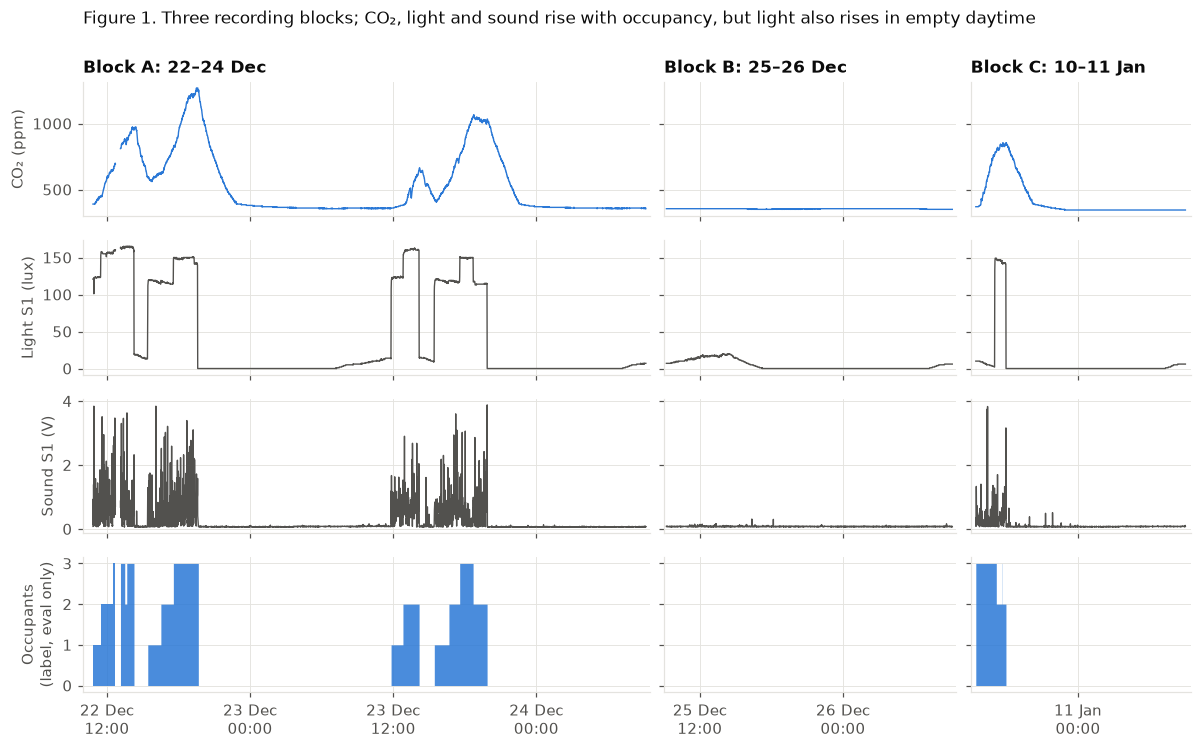

In [4]:
blocks = [(pd.Timestamp("2017-12-22 10:00"), pd.Timestamp("2017-12-24 09:30"), "Block A: 22–24 Dec"),
          (pd.Timestamp("2017-12-25 09:00"), pd.Timestamp("2017-12-26 09:30"), "Block B: 25–26 Dec"),
          (pd.Timestamp("2018-01-10 15:00"), pd.Timestamp("2018-01-11 09:30"), "Block C: 10–11 Jan")]
rows = [("S5_CO2", "CO₂ (ppm)"), ("S1_Light", "Light S1 (lux)"), ("S1_Sound", "Sound S1 (V)"), (LABEL, "Occupants\n(label, eval only)")]
widths = [(b - a).total_seconds() for a, b, _ in blocks]
fig, axes = plt.subplots(len(rows), 3, figsize=(13, 7.2), sharey="row", gridspec_kw={"width_ratios": widths, "wspace": 0.04, "hspace": 0.18})
for j, (a, b, title) in enumerate(blocks):
    for i, (col, lab) in enumerate(rows):
        ax = axes[i, j]
        for _, g in df[(df.ts >= a) & (df.ts <= b)].groupby("segment"):
            if col == LABEL:
                ax.fill_between(g.ts, g[col], step="post", color=C_BLUE, alpha=0.85, linewidth=0)
            else:
                ax.plot(g.ts, g[col], color=C_BLUE if col == "S5_CO2" else INK2, linewidth=0.9)
        ax.set_xlim(a, b)
        if j == 0: ax.set_ylabel(lab)
        if i == 0: ax.set_title(title)
        ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
        if i < len(rows) - 1: ax.tick_params(labelbottom=False)
axes[-1, 0].set_yticks([0, 1, 2, 3])
fig.suptitle("Figure 1. Three recording blocks; CO₂, light and sound rise with occupancy, but light also rises in empty daytime", x=0.125, ha="left", fontsize=11, y=0.97)
fig.savefig(f"{FIG_DIR}/fig1_timeline.png"); plt.show()

**Finding:** the "4 days" are really **three recording blocks** (22–24 Dec, 25–26 Dec, 10–11 Jan), separated by gaps of 24 hours and 15 days. A 25-minute gap on 22 Dec splits the first block in two. Only segments 0, 1 and 3 contain occupancy, and the 25–26 Dec block is entirely empty. Short gaps (≤ 3.6 min) are kept inside segments; windows with too few readings are dropped.

## 1.4 Data Quality and Sensor Behaviour

Sensor data may contain irregularities, unexpected readings or changes in measurement behaviour that affect the interpretation of the investigation.

This subsection examines the quality and behaviour of the available sensor measurements.

The analysis considers missing values, duplicate observations, recording gaps, sensor variation and potential inconsistencies between sensor readings and the occupancy labels.

Particular attention is given to distinguishing unusual environmental conditions from potential data-quality problems.

Importantly, an unusual reading does not automatically indicate a faulty sensor. Its interpretation must consider the surrounding measurements, temporal context and behaviour of other sensors.

In [5]:
# SENSOR DATA QUALITY AND BEHAVIOUR ANALYSIS

# Separate empty and occupied observations for descriptive analysis.
# Occupancy labels are used only to characterise sensor behaviour.
empty_mask = df[LABEL].eq(0)
occupied_mask = df[LABEL].eq(1)

# Sensor measurement characteristics

def get_smallest_increment(series):
    """Return the smallest positive difference between unique readings."""
    values = np.sort(series.dropna().unique())

    if len(values) < 2:
        return np.nan

    differences = np.diff(values)
    positive_differences = differences[differences > 0]

    return positive_differences.min() if len(positive_differences) else np.nan


def get_longest_constant_run(series):
    """Return the longest consecutive run of identical readings."""
    run_groups = series.ne(series.shift()).cumsum()
    return int(series.groupby(run_groups).size().max())


sensor_quality = []

for sensor in SENSORS:
    sensor_quality.append({
        "Sensor": sensor,
        "Unique readings": df[sensor].nunique(),
        "Smallest observed increment": get_smallest_increment(df[sensor]),
        "Longest unchanged run (readings)": get_longest_constant_run(df[sensor])
    })

sensor_quality_df = pd.DataFrame(sensor_quality)

display(
    sensor_quality_df.style
    .format({
        "Smallest observed increment": "{:.3f}",
        "Longest unchanged run (readings)": "{:.0f}"
    }, na_rep="N/A")
    .hide(axis="index")
)

Sensor,Unique readings,Smallest observed increment,Longest unchanged run (readings)
S1_Temp,24,0.060,103
S2_Temp,69,0.060,268
S3_Temp,29,0.060,108
S4_Temp,27,0.060,59
S1_Light,68,1.000,1626
S2_Light,82,1.000,1624
S3_Light,177,1.000,1521
S4_Light,75,1.000,1523
S1_Sound,231,0.010,31
S2_Sound,185,0.010,49


In [6]:
# CO2 baseline across recording segments

co2_baseline_df = (
    df.groupby("segment")["S5_CO2"]
    .agg(
        readings="count",
        median="median",
        lower_baseline=lambda x: x.quantile(0.05),
        upper_baseline=lambda x: x.quantile(0.95)
    )
    .reset_index()
    .rename(columns={
        "segment": "Recording segment",
        "median": "Median CO2 (ppm)",
        "lower_baseline": "5th percentile (ppm)",
        "upper_baseline": "95th percentile (ppm)"
    })
)

display(
    co2_baseline_df.style
    .format({
        "Median CO2 (ppm)": "{:.1f}",
        "5th percentile (ppm)": "{:.1f}",
        "95th percentile (ppm)": "{:.1f}"
    })
    .hide(axis="index")
)

Recording segment,readings,Median CO2 (ppm),5th percentile (ppm),95th percentile (ppm)
0,216,527.5,390.0,675.0
1,5089,375.0,355.0,1035.0
2,2779,355.0,350.0,355.0
3,2045,345.0,345.0,805.0


In [7]:
# Sensor behaviour under empty and occupied conditions

sensor_groups = {
    "Temperature": TEMP,
    "Light": LIGHT,
    "Sound": SOUND,
    "CO2": ["S5_CO2"],
    "Motion (PIR)": PIR
}

occupancy_summary = []

for group_name, sensors in sensor_groups.items():
    for sensor in sensors:

        empty_values = df.loc[empty_mask, sensor]
        occupied_values = df.loc[occupied_mask, sensor]

        occupancy_summary.append({
            "Sensor group": group_name,
            "Sensor": sensor,
            "Empty median": empty_values.median(),
            "Occupied median": occupied_values.median(),
            "Empty readings above zero (%)": (
                (empty_values > 0).mean() * 100
                if group_name in ("Light", "Motion (PIR)")
                else np.nan
            )
        })

occupancy_summary_df = pd.DataFrame(occupancy_summary)

display(
    occupancy_summary_df.style
    .format({
        "Empty median": "{:.2f}",
        "Occupied median": "{:.2f}",
        "Empty readings above zero (%)": "{:.1f}%"
    }, na_rep="—")
    .hide(axis="index")
)

Sensor group,Sensor,Empty median,Occupied median,Empty readings above zero (%)
Temperature,S1_Temp,25.31,25.88,—
Temperature,S2_Temp,25.31,25.75,—
Temperature,S3_Temp,24.88,25.50,—
Temperature,S4_Temp,25.69,26.25,—
Light,S1_Light,0.00,120.00,29.0%
Light,S2_Light,0.00,33.00,29.0%
Light,S3_Light,0.00,58.00,32.1%
Light,S4_Light,0.00,40.00,32.0%
Sound,S1_Sound,0.07,0.26,—
Sound,S2_Sound,0.05,0.09,—


In [8]:

# Hourly occupancy and light statistics

hour = df["ts"].dt.hour
light_positive = df[LIGHT].gt(0).any(axis=1)

hourly_data = pd.DataFrame({
    "hour": hour,
    "occupied": occupied_mask.astype(int),
    "empty": empty_mask.astype(int),
    "empty_with_light": (empty_mask & light_positive).astype(int)
})

# Summarise sensor readings by hour
hourly_summary = (
    hourly_data.groupby("hour")
    .agg(
        total_readings=("occupied", "size"),
        occupied_readings=("occupied", "sum"),
        empty_readings=("empty", "sum"),
        empty_light_positive=("empty_with_light", "sum")
    )
    .reindex(range(24))
)

# Calculate hourly percentages
hourly_summary["occupied_pct"] = (
    hourly_summary["occupied_readings"]
    / hourly_summary["total_readings"] * 100
)

hourly_summary["empty_light_positive_pct"] = (
    hourly_summary["empty_light_positive"]
    / hourly_summary["empty_readings"].replace(0, np.nan) * 100
)

display(hourly_summary.round(1))


,total_readings,occupied_readings,empty_readings,empty_light_positive,occupied_pct,empty_light_positive_pct
hour,,,,,,
0,460,0,460,0,0.0,0.0
1,465,0,465,0,0.0,0.0
2,465,0,465,0,0.0,0.0
3,464,0,464,0,0.0,0.0
4,465,0,465,0,0.0,0.0
5,465,0,465,0,0.0,0.0
6,464,0,464,73,0.0,15.7
7,463,0,463,463,0.0,100.0
8,464,0,464,464,0.0,100.0


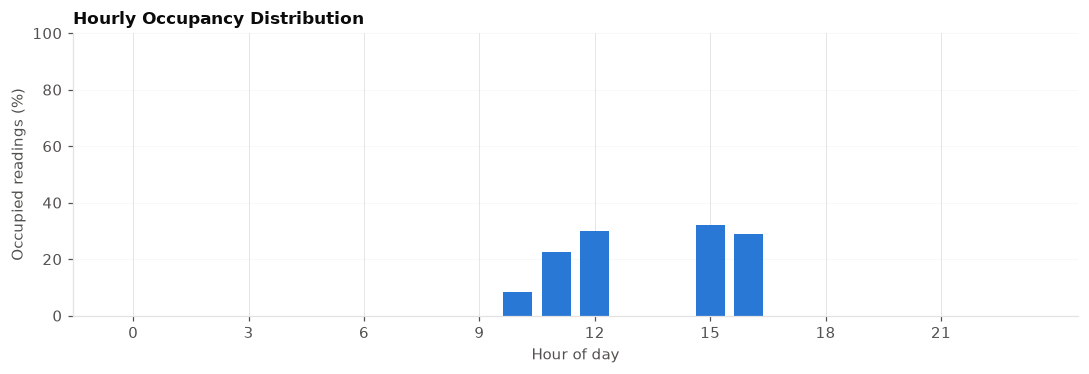

In [9]:
# Percentage of readings labelled as occupied by hour

fig, ax = plt.subplots(figsize=(10, 3.5))

ax.bar(
    hourly_summary.index,
    hourly_summary["occupied_pct"],
    color=C_BLUE,
    width=0.75
)

ax.set_title("Hourly Occupancy Distribution")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Occupied readings (%)")
ax.set_xticks(range(0, 24, 3))
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


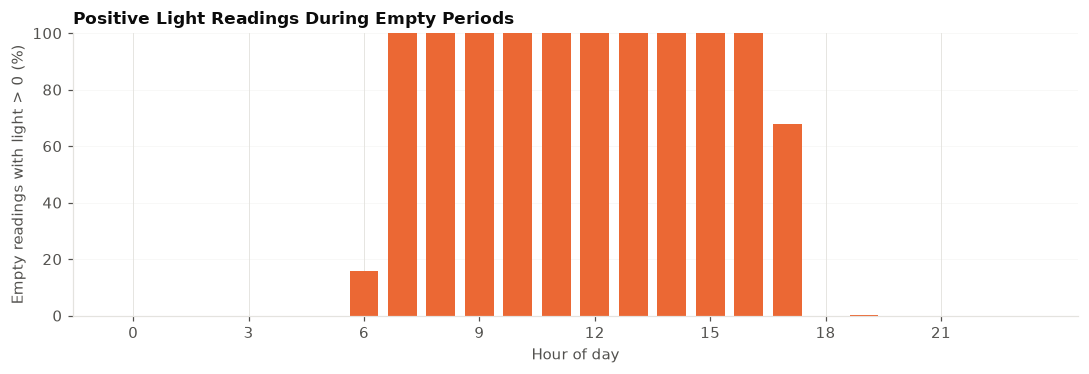

In [10]:

# Percentage of empty readings with positive light measurements by hour

fig, ax = plt.subplots(figsize=(10, 3.5))

ax.bar(
    hourly_summary.index,
    hourly_summary["empty_light_positive_pct"],
    color=C_ORANGE,
    width=0.75
)

ax.set_title("Positive Light Readings During Empty Periods")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Empty readings with light > 0 (%)")
ax.set_xticks(range(0, 24, 3))
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## 1.5 Representation Using Five-Minute Windows

The original dataset contains sensor measurements recorded at approximately 30-second intervals.

For the main data-mining investigation, these readings are transformed into non-overlapping five-minute windows within continuous recording segments.

Each window represents one analytical observation and summarises the sensor behaviour during that period.

The window-based representation provides a more manageable description of room conditions while reducing the influence of highly frequent and potentially noisy measurements.

Sensor-specific summary features are extracted to represent temperature, light, sound, CO₂ and motion behaviour.

The original 30-second measurements are retained separately because aggregating readings into five-minute windows may reduce the temporal detail required to investigate possible room-entry and exit events.

**Analytical object:** Each five-minute window is treated as one observation for the main clustering and anomaly-detection investigation.

In [11]:
FEATURE_GROUPS = {
    "temperature": [f"{c}_mean" for c in TEMP] + [f"{c}_delta" for c in TEMP],
    "light":       [f"{c}_mean" for c in LIGHT],
    "sound":       [f"{c}_mean" for c in SOUND] + [f"{c}_max" for c in SOUND],
    "co2":         ["CO2_excess_mean", "CO2_slope_mean"],
    "motion":      [f"{c}_frac" for c in PIR],
}
NODE_FEATURES = sum(FEATURE_GROUPS.values(), [])
TYPE_FEATURES = ["temp_mean", "temp_delta", "light_mean", "sound_mean", "sound_max", "CO2_excess_mean", "CO2_slope_mean", "pir_frac"]

def make_windows(d, minutes=WINDOW_MIN, min_fill=MIN_FILL):
    # Aggregate 30 s readings into non-overlapping windows inside each contiguous segment.
    d = d.copy()
    d["co2_excess"] = d["S5_CO2"] - d.groupby("segment")["S5_CO2"].transform(lambda s: s.quantile(0.05))
    seg_start = d.groupby("segment")["ts"].transform("min")
    d["win"] = ((d["ts"] - seg_start).dt.total_seconds() // (minutes * 60)).astype(int)
    g = d.groupby(["segment", "win"])
    out = pd.DataFrame({"start": g["ts"].min(), "n_readings": g.size()})
    for c in TEMP:
        out[f"{c}_mean"] = g[c].mean(); out[f"{c}_delta"] = g[c].last() - g[c].first()
    for c in LIGHT: out[f"{c}_mean"] = g[c].mean()
    for c in SOUND: out[f"{c}_mean"] = g[c].mean(); out[f"{c}_max"] = g[c].max()
    out["CO2_excess_mean"] = g["co2_excess"].mean(); out["CO2_slope_mean"] = g["S5_CO2_Slope"].mean()
    for c in PIR: out[f"{c}_frac"] = g[c].mean()
    # sensor-type (node-averaged) representation
    out["temp_mean"]  = out[[f"{c}_mean" for c in TEMP]].mean(axis=1)
    out["temp_delta"] = out[[f"{c}_delta" for c in TEMP]].mean(axis=1)
    out["light_mean"] = out[[f"{c}_mean" for c in LIGHT]].mean(axis=1)
    out["sound_mean"] = out[[f"{c}_mean" for c in SOUND]].mean(axis=1)
    out["sound_max"]  = out[[f"{c}_max" for c in SOUND]].max(axis=1)
    out["pir_frac"]   = out[[f"{c}_frac" for c in PIR]].mean(axis=1)
    # labels: kept in a SEPARATE frame, evaluation only
    lab = pd.DataFrame({"occ_mean": g[LABEL].mean(), "occ_max": g[LABEL].max(),
                        "occ_mode": g[LABEL].agg(lambda s: s.mode().iloc[0]),
                        "transition": g[LABEL].nunique() > 1})
    lab["occupied"] = lab["occ_max"] > 0
    keep = out["n_readings"] >= min_fill * minutes * 2
    out, lab = out[keep].reset_index(), lab[keep].reset_index(drop=True)
    out["date"] = out["start"].dt.date.astype(str); out["hour"] = out["start"].dt.hour
    return out, lab

print("Lag-1 autocorrelation at 30 s:", {c: round(df[c].autocorr(1), 2) for c in ["S1_Temp", "S1_Light", "S5_CO2", "S1_Sound", "S2_Sound", "S6_PIR", "S7_PIR"]})
W, W_lab = make_windows(df)
print(f"{len(W):,} windows of {WINDOW_MIN} min | occupied: {W_lab.occupied.mean():.1%} | windows containing an arrival/departure: {W_lab.transition.mean():.1%}")
print(f"node-level features: {len(NODE_FEATURES)} | sensor-type features: {len(TYPE_FEATURES)}")
W.head()

Lag-1 autocorrelation at 30 s: {'S1_Temp': np.float64(1.0), 'S1_Light': np.float64(1.0), 'S5_CO2': np.float64(1.0), 'S1_Sound': np.float64(0.49), 'S2_Sound': np.float64(0.55), 'S6_PIR': np.float64(0.6), 'S7_PIR': np.float64(0.74)}
1,044 windows of 5 min | occupied: 19.0% | windows containing an arrival/departure: 1.9%
node-level features: 24 | sensor-type features: 8


,segment,win,start,n_readings,S1_Temp_mean,S1_Temp_delta,S2_Temp_mean,S2_Temp_delta,S3_Temp_mean,S3_Temp_delta,...,S6_PIR_frac,S7_PIR_frac,temp_mean,temp_delta,light_mean,sound_mean,sound_max,pir_frac,date,hour
0,0,0,2017-12-22 10:49:41,10,24.988000,0.06,24.774000,0.06,24.554,0.00,...,0.200000,0.1,24.940500,0.0600,61.950000,0.29300,3.84,0.150000,2017-12-22,10
1,0,1,2017-12-22 10:54:47,10,25.060000,0.00,24.845000,0.07,24.616,0.07,...,0.800000,0.1,25.012750,0.0500,64.775000,0.24075,2.20,0.450000,2017-12-22,10
2,0,2,2017-12-22 10:59:54,10,25.123000,0.00,24.880000,0.00,24.660,0.06,...,0.500000,0.0,25.049750,0.0300,65.175000,0.21400,1.57,0.250000,2017-12-22,10
3,0,3,2017-12-22 11:05:00,10,25.190000,0.00,24.892000,0.06,24.690,0.00,...,0.100000,0.0,25.089750,0.0150,64.925000,0.11250,0.93,0.050000,2017-12-22,11
4,0,4,2017-12-22 11:10:06,9,25.203333,0.06,24.933333,0.00,24.730,0.00,...,0.222222,0.0,25.122222,0.0325,65.972222,0.22750,1.44,0.111111,2017-12-22,11


### Transformation and scaling
Distance-based clustering and anomaly methods (k-means, GMM, LOF, DBSCAN) are dominated by whichever feature has the largest numeric range. Light and sound are heavily right-skewed with many zeros, so they get a `log1p` transform, then **every feature is standardised** (z-scores).

For discovery, the scaler is fit on all windows, which is fine because no labels are involved. **For any predictive extension, refit the scaler on the training days only** using `scale_features(train, test)`.

In [12]:
LOG_COLS = [c for c in NODE_FEATURES + TYPE_FEATURES if any(k in c for k in ("Light", "light", "Sound", "sound"))]

def transform(Wdf, cols):
    X = Wdf[cols].copy()
    for c in set(cols) & set(LOG_COLS): X[c] = np.log1p(X[c])
    return X

def scale_features(train, test=None, cols=NODE_FEATURES):
    # log1p skewed columns, then z-score using statistics from `train` only.
    sc = StandardScaler().fit(transform(train, cols))
    Xtr = pd.DataFrame(sc.transform(transform(train, cols)), columns=cols, index=train.index)
    if test is None: return Xtr
    return Xtr, pd.DataFrame(sc.transform(transform(test, cols)), columns=cols, index=test.index)

X_node = scale_features(W, cols=NODE_FEATURES)
X_type = scale_features(W, cols=TYPE_FEATURES)
X_node.describe().loc[["mean", "std"]].round(2)

,S1_Temp_mean,S2_Temp_mean,S3_Temp_mean,S4_Temp_mean,S1_Temp_delta,S2_Temp_delta,S3_Temp_delta,S4_Temp_delta,S1_Light_mean,S2_Light_mean,...,S3_Sound_mean,S4_Sound_mean,S1_Sound_max,S2_Sound_max,S3_Sound_max,S4_Sound_max,CO2_excess_mean,CO2_slope_mean,S6_PIR_frac,S7_PIR_frac
mean,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,...,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 1.7 How Preparation Choices Influence the Analysis

Data preparation is not simply a preliminary cleaning step. It influences how observations are compared and, consequently, the patterns and unusual observations that can be discovered.

This subsection examines the implications of important preparation decisions, including feature scaling and the choice of time-window duration.

The analysis considers the trade-off between retaining detailed temporal information and creating more stable observations for data mining.

These comparisons help establish whether the selected representation is appropriate for the investigation and identify limitations that should be considered when interpreting subsequent results.

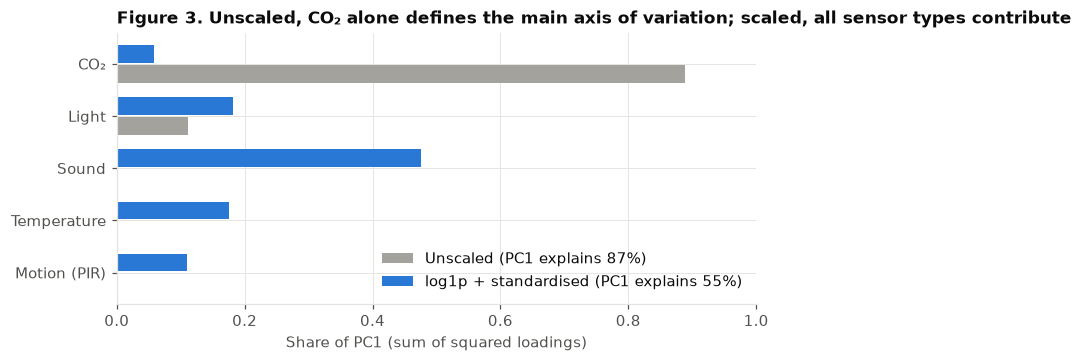

,unscaled,log1p + standardised
co2,0.888,0.059
light,0.112,0.182
sound,0.000,0.476
temperature,0.000,0.175
motion,0.000,0.109


In [13]:
def pc1_share_by_group(X, cols):
    p = PCA(n_components=1, random_state=RANDOM_SEED).fit(X)
    load = pd.Series(np.abs(p.components_[0]) ** 2, index=cols)  # squared loadings sum to 1
    grp = {c: g for g, cs in FEATURE_GROUPS.items() for c in cs}
    return load.groupby(grp).sum(), p.explained_variance_ratio_[0]

raw_share, raw_ev = pc1_share_by_group(W[NODE_FEATURES], NODE_FEATURES)
sc_share,  sc_ev  = pc1_share_by_group(X_node, NODE_FEATURES)
order = ["co2", "light", "sound", "temperature", "motion"]
comp = pd.DataFrame({"unscaled": raw_share, "log1p + standardised": sc_share}).loc[order]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
yy = np.arange(len(order)); h = 0.38
ax.barh(yy + h/2, comp["unscaled"], height=h - 0.04, color=C_GREY, label=f"Unscaled (PC1 explains {raw_ev:.0%})")
ax.barh(yy - h/2, comp["log1p + standardised"], height=h - 0.04, color=C_BLUE, label=f"log1p + standardised (PC1 explains {sc_ev:.0%})")
ax.set_yticks(yy); ax.set_yticklabels(["CO₂", "Light", "Sound", "Temperature", "Motion (PIR)"]); ax.invert_yaxis()
ax.set_xlabel("Share of PC1 (sum of squared loadings)"); ax.set_xlim(0, 1)
ax.legend(loc="lower right")
ax.set_title("Figure 3. Unscaled, CO₂ alone defines the main axis of variation; scaled, all sensor types contribute")
fig.savefig(f"{FIG_DIR}/fig3_scaling_effect.png"); plt.show()
comp.round(3)

In [14]:

# Evaluate different aggregation window lengths

window_lengths = [1, 2, 5, 10, 15, 30]
window_results = []

for minutes in window_lengths:
    windows, labels = make_windows(df, minutes=minutes)

    sound_autocorr = windows["S1_Sound_mean"].autocorr(lag=1)

    window_results.append({
        "window (min)": minutes,
        "windows": len(windows),
        "% windows mixing an arrival/departure": (
            100 * labels["transition"].mean()
        ),
        "lag-1 autocorr of S1 sound": sound_autocorr
    })

wl = pd.DataFrame(window_results).set_index("window (min)")


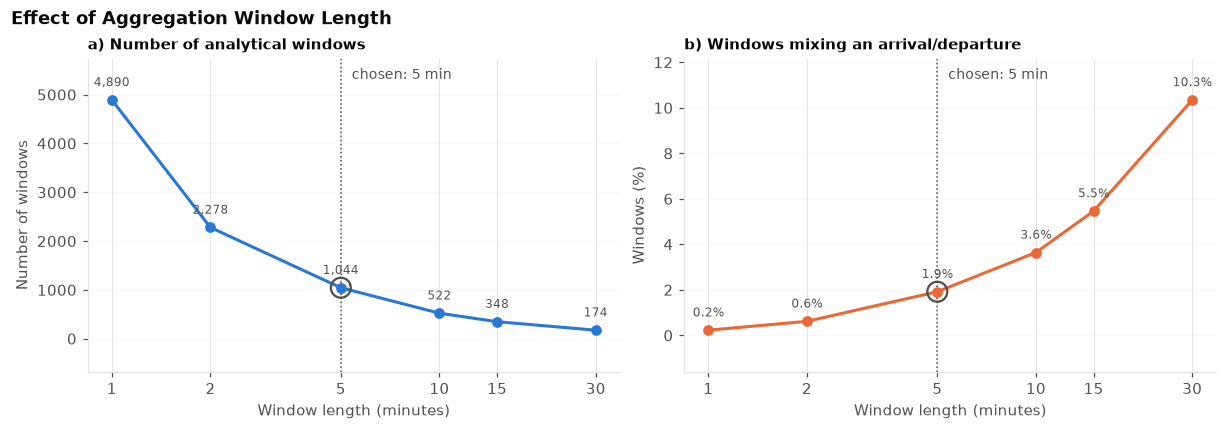

In [15]:
from matplotlib.ticker import ScalarFormatter

# Visualise the effect of aggregation window length
pct_col = "% windows mixing an arrival/departure"

fig, axes = plt.subplots(
    1, 2, figsize=(11, 3.8), sharex=True, constrained_layout=True
)

panels = [
    (axes[0], "windows", C_BLUE,
     "a) Number of analytical windows", "Number of windows", "{:,.0f}"),
    (axes[1], pct_col, C_ORANGE,
     "b) Windows mixing an arrival/departure", "Windows (%)", "{:.1f}%"),
]

for ax, col, color, title, ylabel, fmt in panels:
    # Main line
    ax.plot(wl.index, wl[col], marker="o", markersize=6,
            linewidth=2, color=color, zorder=3)

    # Value label on every point
    for x, v in wl[col].items():
        ax.annotate(fmt.format(v), (x, v), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=8, color=INK2)

    # Highlight the chosen window with a ring
    ax.scatter(WINDOW_MIN, wl.loc[WINDOW_MIN, col], s=170,
               facecolors="none", edgecolors=INK2, linewidths=1.5, zorder=4)

    # Reference line and label for the chosen window
    ax.axvline(WINDOW_MIN, color=INK2, linestyle=":", linewidth=1)
    ax.text(WINDOW_MIN * 1.08, 0.97, f"chosen: {WINDOW_MIN} min",
            transform=ax.get_xaxis_transform(),
            va="top", ha="left", fontsize=9, color=INK2)

    # Log x-axis so 1, 2, 5, 10, 15, 30 are spread out evenly
    ax.set_xscale("log")
    ax.set_xticks(wl.index)
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.minorticks_off()

    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("Window length (minutes)")
    ax.set_ylabel(ylabel)
    ax.margins(y=0.18)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig.suptitle("Effect of Aggregation Window Length",
             x=0.0, ha="left", fontsize=12, fontweight="bold")

fig.savefig(f"{FIG_DIR}/fig4_window_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:

# Compare window lengths numerically

display(wl.round(3))


,windows,% windows mixing an arrival/departure,lag-1 autocorr of S1 sound
window (min),,,
1,4890,0.225,0.647
2,2278,0.615,0.738
5,1044,1.916,0.798
10,522,3.640,0.840
15,348,5.460,0.816
30,174,10.345,0.817


## 1.8 Exporting Prepared Data for Subsequent Analysis

The prepared datasets and feature representations are exported for use in the subsequent stages of the group investigation.

These outputs provide a consistent foundation for clustering, sensor-representation comparisons, anomaly detection and temporal analysis.

The occupancy labels are maintained separately from the unsupervised feature inputs so that they can be used for evaluation and interpretation without influencing the discovery process.

The exported data also support reproducibility and consistency across the different analytical contributions of the group.

In [17]:

# 1.8 Exporting Prepared Data for Subsequent Analysis

from pathlib import Path
import json

# Ensure the output directory exists.
OUT_DIR = Path(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Export original sensor readings.
df.to_csv(OUT_DIR / "points_30s.csv", index=False)

# Export five-minute aggregated sensor features.
W.to_csv(OUT_DIR / "windows_5min.csv", index=False)

# Export occupancy labels separately for evaluation.
W_lab.to_csv(OUT_DIR / "windows_5min_labels.csv", index=False)

# Export scaled feature representations.
X_node.to_csv(OUT_DIR / "X_node_scaled.csv", index=False)
X_type.to_csv(OUT_DIR / "X_type_scaled.csv", index=False)

# Export feature-group definitions.
with open(OUT_DIR / "feature_groups.json", "w") as f:
    json.dump(
        {
            "node_level": FEATURE_GROUPS,
            "sensor_type_level": TYPE_FEATURES
        },
        f,
        indent=2
    )

# Verify exported files.
print("Exported files:")
for file in sorted(OUT_DIR.iterdir()):
    if file.is_file():
        print(f"  {file.name}")

print("\nWindows per date:")
print(W.groupby("date").size().to_dict())


Exported files:
  X_node_scaled.csv
  X_type_scaled.csv
  feature_groups.json
  points_30s.csv
  windows_5min.csv
  windows_5min_labels.csv

Windows per date:
{'2017-12-22': 150, '2017-12-23': 287, '2017-12-24': 109, '2017-12-25': 178, '2017-12-26': 109, '2018-01-10': 103, '2018-01-11': 108}


# 2. Discovering Room-Usage Patterns Through Clustering

Following the preparation of the sensor data, this section investigates whether recurring room-usage patterns can be identified from unlabelled environmental measurements.

Clustering is used to group observations according to similarities in their sensor-derived features. The objective is to determine whether the room exhibits distinct patterns of environmental and activity-related behaviour.

The analysis focuses on the structure of the prepared five-minute observations rather than using occupancy labels to determine cluster membership.

The discovered groups are subsequently examined to understand their sensor characteristics, temporal distribution and potential interpretation in the context of room usage.

The existence of a cluster does not automatically establish a particular occupancy state. Interpretation is based on the observed sensor characteristics and supporting evidence.

## 2.1 Clustering Objective and Analytical Representation

The purpose of clustering is to investigate whether the prepared sensor observations contain distinct and recurring patterns of room conditions and activity.

The analytical unit is one **five-minute observation window**. Each window is represented by sensor-derived features describing environmental conditions, including temperature, light, sound, CO₂ and passive infrared (PIR) motion measurements.

The clustering input is constructed using the prepared and scaled feature representation (`X_node`). Scaling is important because the sensor features have different measurement ranges. Without scaling, features with larger numerical values could have a disproportionate influence on the clustering results.

Occupancy labels are deliberately excluded from the clustering input. This ensures that the groups are discovered from the sensor measurements rather than being determined by the known occupancy information. The occupancy labels are retained separately for subsequent evaluation and interpretation.

A meaningful cluster should contain observations with similar sensor characteristics. By examining the sensor profiles and temporal distribution of each group, we aim to identify recurring room conditions and investigate what they may indicate about room usage.

However, similarity in sensor measurements does not necessarily confirm a particular occupancy state. Cluster interpretations must therefore consider the available evidence and the limitations of the sensors.

In [18]:
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

In [19]:
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

Xc = X_node.values   # the matrix we cluster (no labels)

def hopkins(X, frac=0.1, seed=0):
    rng = np.random.default_rng(seed)
    n = len(X); m = int(frac * n)                       # use 10% of windows
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    # w: real windows -> nearest OTHER real window (column 1, because column 0 is itself)
    w = nn.kneighbors(X[rng.choice(n, m, replace=False)])[0][:, 1]
    # u: random points spread over the same range -> nearest real window
    fake = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, X.shape[1]))
    u = nn.kneighbors(fake, n_neighbors=1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())                                           # write the formula

H = np.array([hopkins(Xc, seed=s) for s in range(10)])  # repeat 10 times
print(f"Hopkins: mean {H.mean():.3f}, sd {H.std():.3f}")     # print the mean

Hopkins: mean 0.901, sd 0.011



#### Interpretation

The Hopkins Statistic provides an initial indication of whether the sensor measurements contain natural grouping patterns.

A result closer to 1 indicates that the observations are more clustered than would be expected from randomly distributed data.

This supports our decision to investigate clustering further using K-Means.

However, Hopkins alone does not prove that the final clusters are meaningful. We therefore use additional evaluation measures when selecting the number of clusters.


## 2.2 Clustering Methodology

We use **K-Means clustering** to investigate the structure of the prepared sensor observations. K-Means is an unsupervised learning algorithm that groups observations according to their similarity in the feature space.

The algorithm works by assigning each observation to the nearest cluster centre, also known as a centroid. The centroids are updated iteratively to minimise the within-cluster sum of squares (WSS), which measures the variation between observations and their assigned cluster centres.

In this investigation, K-Means uses the prepared and scaled sensor features from `X_node`. Euclidean distance is used to measure the similarity between observations. Since the features have been standardised, no single sensor measurement should dominate the distance calculation simply because it has a larger numerical scale.

K-Means is suitable for this initial investigation because it provides a straightforward way to identify groups of observations with similar sensor characteristics. However, it has limitations. The algorithm requires the number of clusters to be specified in advance and can be influenced by outliers, initial centroid positions and the shape of the underlying data. It may also represent irregularly shaped groups less effectively.

Before selecting the final number of clusters, we first examine whether the dataset shows evidence of natural grouping using the Hopkins Statistic. We then compare different values of K using multiple evaluation measures, including:

- **Within-Cluster Sum of Squares (WSS):** Measures the variation within clusters and helps identify an appropriate number of clusters.
- **Silhouette Score:** Evaluates how well observations fit within their assigned clusters compared with other clusters.
- **Davies–Bouldin Index:** Measures the similarity between clusters, with lower values generally indicating better separation.
- **Clustering Stability:** Uses repeated subsamples and the Adjusted Rand Index (ARI) to examine whether similar groupings are produced when the data sample changes.

These measures are considered together because no single metric is sufficient to establish that a clustering solution is meaningful. The final choice should balance cluster separation, stability, cluster size and interpretability in the context of room usage.

In [20]:
K_RANGE = range(2, 9)
rng = np.random.default_rng(RANDOM_SEED)
results = []

for k in K_RANGE:
    # 1. fit k-means on all windows
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_SEED).fit(Xc)

    # 2. stability: refit on 20 random 80% samples, compare with the full fit using ARI
    boot = []
    for b in range(20):
        idx = rng.choice(len(Xc), int(0.8 * len(Xc)), replace=False)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Xc[idx])
        boot.append(adjusted_rand_score(km.labels_, km_b.predict(Xc)))

    # 3. store the scores
    results.append({"k": k,
                    "WSS": km.inertia_,
                    "silhouette": silhouette_score(Xc, km.labels_),
                    "Davies-Bouldin": davies_bouldin_score(Xc, km.labels_),
                    "stability (mean ARI)": np.mean(boot),
                    "stability sd": np.std(boot),
                    "smallest cluster": np.bincount(km.labels_).min()})

ksel = pd.DataFrame(results).set_index("k")
ksel.round(3)

,WSS,silhouette,Davies-Bouldin,stability (mean ARI),stability sd,smallest cluster
k,,,,,,
2,13884.657,0.554,0.967,0.979,0.014,181
3,11679.406,0.320,1.341,0.948,0.098,152
4,10254.357,0.293,1.390,0.977,0.022,99
5,9127.432,0.309,1.356,0.987,0.007,82
6,8535.694,0.314,1.436,0.979,0.009,24
7,8125.884,0.293,1.320,0.921,0.037,5
8,7723.774,0.304,1.468,0.838,0.156,5


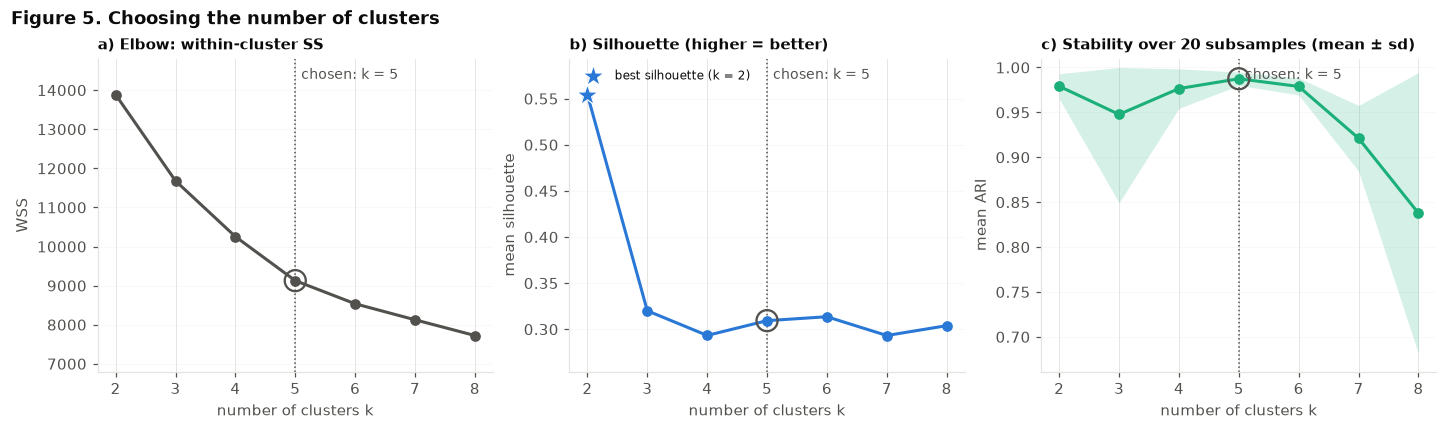

In [21]:
# Set this to the k you actually chose
K_CHOSEN = 5  # <- change to your selected k

k_vals = ksel.index.to_numpy()
best_sil_k = ksel["silhouette"].idxmax()

ari = ksel["stability (mean ARI)"]
ari_sd = ksel["stability sd"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)

# a) Elbow
ax = axes[0]
ax.plot(k_vals, ksel["WSS"], marker="o", markersize=6, linewidth=2, color=INK2, zorder=3)
ax.set_title("a) Elbow: within-cluster SS", loc="left", fontsize=10)
ax.set_ylabel("WSS")

# b) Silhouette
ax = axes[1]
ax.plot(k_vals, ksel["silhouette"], marker="o", markersize=6, linewidth=2, color=C_BLUE, zorder=3)
ax.scatter(best_sil_k, ksel.loc[best_sil_k, "silhouette"], marker="*", s=220,
           color=C_BLUE, edgecolors="white", linewidths=0.8, zorder=5,
           label=f"best silhouette (k = {best_sil_k})")
ax.legend(loc="best", frameon=False, fontsize=8)
ax.set_title("b) Silhouette (higher = better)", loc="left", fontsize=10)
ax.set_ylabel("mean silhouette")

# c) Stability: line with an sd band instead of error bars
ax = axes[2]
ax.plot(k_vals, ari, marker="o", markersize=6, linewidth=2, color=C_AQUA, zorder=3)
ax.fill_between(k_vals, ari - ari_sd, np.minimum(ari + ari_sd, 1.0),
                color=C_AQUA, alpha=0.18, linewidth=0)
ax.set_ylim(min(0.8, (ari - ari_sd).min() - 0.02), 1.01)
ax.set_title("c) Stability over 20 subsamples (mean ± sd)", loc="left", fontsize=10)
ax.set_ylabel("mean ARI")

# Shared formatting
panel_cols = ["WSS", "silhouette", "stability (mean ARI)"]
for ax, col in zip(axes, panel_cols):
    # Highlight the chosen k
    ax.axvline(K_CHOSEN, color=INK2, linestyle=":", linewidth=1, zorder=1)
    ax.scatter(K_CHOSEN, ksel.loc[K_CHOSEN, col], s=190, facecolors="none",
               edgecolors=INK2, linewidths=1.5, zorder=4)
    ax.text(K_CHOSEN + 0.1, 0.97, f"chosen: k = {K_CHOSEN}",
            transform=ax.get_xaxis_transform(), va="top", ha="left",
            fontsize=9, color=INK2)

    ax.set_xlabel("number of clusters k")
    ax.set_xticks(list(K_RANGE))
    ax.margins(y=0.15)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig.suptitle("Figure 5. Choosing the number of clusters",
             x=0.0, ha="left", fontsize=12, fontweight="bold")

fig.savefig(f"{FIG_DIR}/fig5_choose_k.png", dpi=300, bbox_inches="tight")
plt.show()


#### Interpreting the Cluster Selection Results

Figure 5 compares the performance of K-Means across different values of K (2 to 8).

The three plots help us understand:

- **Elbow plot:** How much the within-cluster variation decreases as more clusters are added.
- **Silhouette plot:** How well the clusters are separated.
- **Stability plot:** Whether similar groups are produced when different subsets of the data are used.

We consider these results together rather than relying on one score alone.

Based on the overall clustering analysis, we select **K = 5** for the final model. This provides five room states that can be investigated and interpreted using their sensor characteristics.


## 2.3 Selecting and Evaluating Cluster Structure

Selecting an appropriate clustering configuration is important because different model settings can produce different groupings.

This subsection examines the evidence used to assess the resulting cluster structure.

The evaluation considers the separation and consistency of the discovered groups, alongside whether the resulting clusters provide an interpretable description of the sensor observations.

Quantitative evaluation is considered together with visual inspection and the practical meaning of the resulting groups.

The final interpretation should reflect the strengths and limitations of the available evidence.

In [22]:
K_FINAL = 5
km_final = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_SEED).fit(Xc)
W["cluster"] = km_final.labels_

# distance of each window to its own cluster centre (useful later for the anomaly person)
W["dist_to_centroid"] = np.linalg.norm(Xc - km_final.cluster_centers_[km_final.labels_], axis=1)

# median raw (unscaled) values per cluster, easier to interpret than z-scores
prof = W.groupby("cluster")[TYPE_FEATURES + ["hour"]].median().round(2)
prof["windows"] = W["cluster"].value_counts().sort_index()
prof

,temp_mean,temp_delta,light_mean,sound_mean,sound_max,CO2_excess_mean,CO2_slope_mean,pir_frac,hour,windows
cluster,,,,,,,,,,
0,26.18,0.01,141.11,0.64,3.32,492.50,1.67,0.57,17.0,82
1,25.28,0.00,0.00,0.06,0.09,5.00,0.00,0.00,5.0,545
2,25.86,-0.03,0.00,0.06,0.08,380.39,-2.12,0.00,19.5,88
3,25.10,0.00,20.27,0.07,0.10,5.00,0.00,0.00,10.0,216
4,25.93,0.01,69.88,0.26,1.28,205.00,0.80,0.28,15.0,113


## 2.4 Interpreting the Discovered Room-Usage Patterns

After identifying the cluster structure, the resulting groups are examined using their sensor characteristics and temporal behaviour.

This subsection investigates how temperature, light, sound, CO₂ and motion measurements vary across the discovered clusters.

The purpose is to understand what distinguishes one group of observations from another and whether the differences represent recurring room-usage patterns.

Occupancy labels may be used as supporting evaluation evidence, but the clusters are interpreted primarily through their sensor-derived characteristics.

The findings from this subsection provide the basis for examining sensor contributions and the robustness of the discovered structure.

In [23]:
# Name each cluster from its sensor profile (labels are NOT used)
def name_cluster(p, busiest):
    if p["pir_frac"] > 0:                       # motion in a typical window -> people present
        return "Busy: high light, CO₂ rising" if p.name == busiest else "Occupied: moderate activity"
    if p["light_mean"] > 0:                     # no motion but light > 0 -> daylight
        return "Empty: daylight only"
    if p["CO2_slope_mean"] < -0.5:              # dark, no motion, CO₂ still falling -> people just left
        return "Recently vacated: dark, CO₂ falling"
    return "Empty: dark (night)"

# of the clusters with motion, the one with the fastest-rising CO₂ is the "busy" one
busiest = prof.loc[prof["pir_frac"] > 0, "CO2_slope_mean"].idxmax()

CLUSTER_NAMES = {c: name_cluster(prof.loc[c], busiest) for c in prof.index}
assert len(set(CLUSTER_NAMES.values())) == K_FINAL, "two clusters got the same name, so check `prof`"

W["cluster_name"] = W["cluster"].map(CLUSTER_NAMES)

# fixed display order for every plot (quiet -> busy)
ORDER = ["Empty: dark (night)", "Empty: daylight only", "Recently vacated: dark, CO₂ falling",
         "Occupied: moderate activity", "Busy: high light, CO₂ rising"]
print(CLUSTER_NAMES)
W["cluster_name"].value_counts().loc[ORDER]

{0: 'Busy: high light, CO₂ rising', 1: 'Empty: dark (night)', 2: 'Recently vacated: dark, CO₂ falling', 3: 'Empty: daylight only', 4: 'Occupied: moderate activity'}


cluster_name
Empty: dark (night)                    545
Empty: daylight only                   216
Recently vacated: dark, CO₂ falling     88
Occupied: moderate activity            113
Busy: high light, CO₂ rising            82
Name: count, dtype: int64

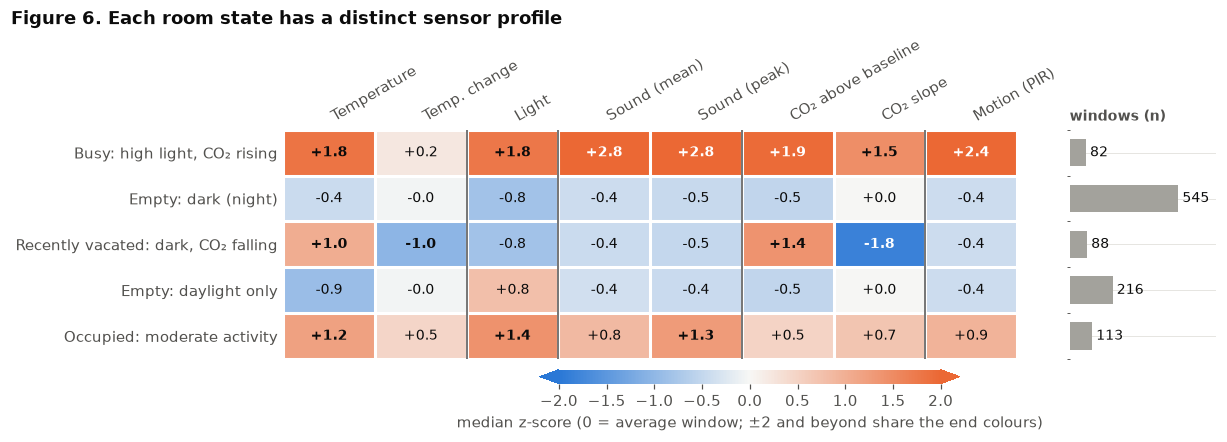

In [24]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

ORDER = list(CLUSTER_NAMES.values())          # row order on the plot
Z = (X_type.assign(cluster_name=W["cluster_name"])
           .groupby("cluster_name").median().loc[ORDER])
counts = W["cluster_name"].value_counts().loc[ORDER]

nice = {"temp_mean": "Temperature", "temp_delta": "Temp. change", "light_mean": "Light",
        "sound_mean": "Sound (mean)", "sound_max": "Sound (peak)",
        "CO2_excess_mean": "CO₂ above baseline", "CO2_slope_mean": "CO₂ slope",
        "pir_frac": "Motion (PIR)"}

# Which sensor each feature belongs to (used for separators between groups)
group = {"temp_mean": "temp", "temp_delta": "temp", "light_mean": "light",
         "sound_mean": "sound", "sound_max": "sound",
         "CO2_excess_mean": "co2", "CO2_slope_mean": "co2", "pir_frac": "pir"}

# Theme: blue (below average) -> near-white (average) -> orange (above average)
cmap = LinearSegmentedColormap.from_list("blue_orange", [C_BLUE, "#F7F7F5", C_ORANGE])
LIM = 2
norm = TwoSlopeNorm(vmin=-LIM, vcenter=0, vmax=LIM)

fig, (ax, axn) = plt.subplots(
    1, 2, figsize=(11, 3.9), sharey=True, constrained_layout=True,
    gridspec_kw={"width_ratios": [1, 0.2]}
)

# --- Heatmap ---
im = ax.imshow(Z.values, cmap=cmap, norm=norm, aspect="auto")

ax.set_xticks(range(Z.shape[1]))
ax.set_xticklabels([nice[c] for c in Z.columns], rotation=30, ha="left")
ax.xaxis.tick_top()
ax.set_yticks(range(len(ORDER)))
ax.set_yticklabels(ORDER)

# White cell borders
ax.set_xticks(np.arange(-0.5, Z.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-0.5, Z.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)

# Thicker separators between sensor groups
cols = list(Z.columns)
for j in range(len(cols) - 1):
    if group[cols[j]] != group[cols[j + 1]]:
        ax.axvline(j + 0.5, color=INK, linewidth=1.2, alpha=0.6)

# Cell values: text colour chosen from cell brightness, bold when |z| >= 1
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        v = Z.values[i, j]
        r, g, b, _ = cmap(norm(v))
        dark_cell = (0.299 * r + 0.587 * g + 0.114 * b) < 0.55
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                fontweight="bold" if abs(v) >= 1 else "normal",
                color="white" if dark_cell else INK)

# --- Cluster size panel ---
axn.barh(range(len(ORDER)), counts.values, color=C_GREY, height=0.6)
for i, n in enumerate(counts.values):
    axn.text(n, i, f" {n:,}", va="center", ha="left", fontsize=9, color=INK)
axn.set_xlim(0, counts.max() * 1.35)
axn.set_xticks([])
axn.tick_params(left=False)
axn.set_title("windows (n)", fontsize=9, color=INK2)
for s in axn.spines.values():
    s.set_visible(False)

# --- Colourbar ---
cb = fig.colorbar(im, ax=[ax, axn], location="bottom", shrink=0.45,
                  pad=0.04, aspect=30, extend="both")
cb.set_label("median z-score (0 = average window; ±2 and beyond share the end colours)")
cb.outline.set_visible(False)

fig.suptitle("Figure 6. Each room state has a distinct sensor profile",
             x=0.0, ha="left", fontsize=12, fontweight="bold")

fig.savefig(f"{FIG_DIR}/fig6_cluster_profiles.png", dpi=300, bbox_inches="tight")
plt.show()


### 2.5 Analysing Room States Over Time

Identifying five clusters is useful, but we also need to understand when these room conditions occur.

In this step, we visualise the cluster assignments across the three recording periods.

Each colour represents one of the five identified room states. We also display the recorded occupancy count underneath the cluster timeline.

The occupancy information is included only for comparison and evaluation. It was not used to train the K-Means model.

#### What are we looking for?

We want to understand whether the identified room states appear in meaningful time periods.

For example:

- Does the empty nighttime cluster appear during overnight periods?
- Does the daylight cluster appear during daytime when the room is empty?
- Does the recently vacated cluster appear after occupied periods?
- Do the occupied clusters appear when people are recorded inside the room?

If the clusters represent meaningful room conditions, we would expect them to form reasonably consistent periods rather than appearing randomly throughout the timeline.


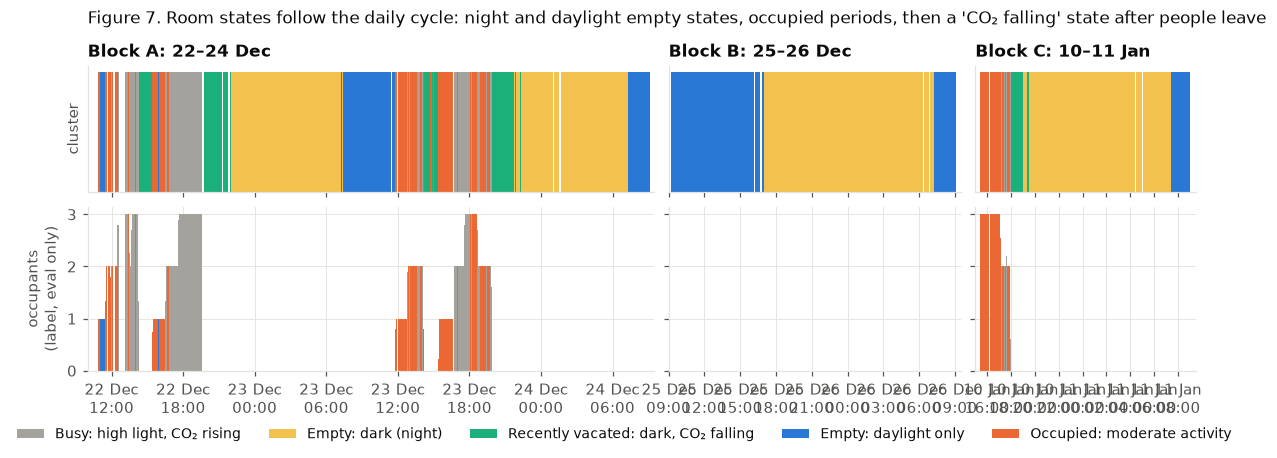

In [25]:
CL_COL = dict(zip(ORDER, [C_GREY, "#f2c14e", C_AQUA, C_BLUE, C_ORANGE]))

fig, axes = plt.subplots(2, 3, figsize=(13, 3.6), sharey="row",
                         gridspec_kw={"width_ratios": widths, "height_ratios": [1, 1.3],
                                      "wspace": 0.04, "hspace": 0.1})
occ = W_lab["occ_mean"]   # evaluation only

for j, (a, b, title) in enumerate(blocks):
    in_block = (W["start"] >= a) & (W["start"] <= b)
    for n in ORDER:
        m = in_block & (W["cluster_name"] == n)
        axes[0, j].bar(W.loc[m, "start"], 1, width=pd.Timedelta(minutes=5), color=CL_COL[n],
                       linewidth=0, align="edge", label=n if j == 0 else None)
        axes[1, j].bar(W.loc[m, "start"], occ[m], width=pd.Timedelta(minutes=5), color=CL_COL[n],
                       linewidth=0, align="edge")
    for ax in axes[:, j]:
        ax.set_xlim(a, b)
        # ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
    axes[0, j].set_title(title); axes[0, j].set_yticks([])
    axes[0, j].tick_params(labelbottom=False); axes[0, j].grid(False)

axes[0, 0].set_ylabel("cluster")
axes[1, 0].set_ylabel("occupants\n(label, eval only)"); axes[1, 0].set_yticks([0, 1, 2, 3])
fig.legend(loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.1), fontsize=9)
fig.suptitle("Figure 7. Room states follow the daily cycle: night and daylight empty states, "
             "occupied periods, then a 'CO₂ falling' state after people leave",
             x=0.125, ha="left", fontsize=11, y=1.02)
fig.savefig(f"{FIG_DIR}/fig7_clusters_timeline.png"); plt.show()


#### Interpretation of the Timeline

Figure 7 shows that the identified room states follow recognisable patterns across the recording periods.

**Key observations:**

1. **Nighttime conditions:** The dark, empty cluster mainly appears overnight, when light and movement measurements are low.

2. **Daylight conditions:** The daylight-only cluster appears during daytime periods, including the Christmas recording block when the room was recorded as empty.

3. **Recently vacated conditions:** The CO₂-falling cluster appears immediately after occupied periods end. This supports the interpretation that CO₂ takes time to decrease after people leave.

4. **Occupied conditions:** The two occupied clusters appear during periods when people are present. They sometimes alternate rapidly because they represent different sensor activity patterns.

These observations suggest that the clustering model is capturing meaningful changes in room conditions over time.

However, the two occupied clusters do not reliably distinguish the exact number of people in the room.



### 2.6 Evaluating the Clustering Results Against Occupancy Labels

After identifying and interpreting the five room states, we evaluate whether they correspond to the actual recorded occupancy information.

This is an important step because our clustering model was trained without using occupancy labels.

We now compare the cluster assignments with `W_lab`, which contains the recorded occupancy information for each 5-minute window.

#### What do we evaluate?

We investigate three main questions:

**1. Can the model distinguish an empty room from an occupied room?**

We combine the two occupied clusters into one category and compare them with the recorded empty/occupied labels.

We calculate the percentage of windows where both agree.

**2. How well do the clusters represent the exact number of occupants?**

We compare the five cluster assignments against the recorded head-count categories (0, 1, 2, and 3 people) using the Adjusted Rand Index (ARI).

**3. How do five clusters relate to a simpler two-cluster solution?**

We also run K-Means with K = 2 to investigate whether the five room states provide additional detail beyond a simple empty-versus-occupied distinction.

#### Understanding the evaluation measures

- **Agreement percentage:** The proportion of windows where the predicted empty/occupied category matches the recorded occupancy category.
- **Adjusted Rand Index (ARI):** Measures the similarity between two groupings while accounting for agreement that could occur by chance. A value closer to 1 indicates stronger agreement, while values around 0 indicate agreement similar to chance.

These comparisons help us understand both the strengths and limitations of the clustering approach.


In [26]:
# 1. How many windows of each head-count fall in each cluster?
ct = pd.crosstab(W["cluster_name"], W_lab["occ_mode"]).loc[ORDER]
ct.columns = [f"{c} people" for c in ct.columns]
print("Windows per cluster by most common head-count:")
display(ct)

# 2. Empty vs occupied: do the two 'people' clusters match the label?
occ_pred = W["cluster_name"].str.startswith(("Busy", "Occupied"))
agree = 100 * (occ_pred == W_lab["occupied"]).mean()
print(f"Empty vs occupied agreement: {agree:.1f}%  "
      f"(ARI {adjusted_rand_score(W_lab['occupied'], occ_pred):.2f})")

# 3. Exact head-count (0, 1, 2, 3): much harder
print(f"ARI, 5 clusters vs head-count 0–3: {adjusted_rand_score(W_lab['occ_mode'], W['cluster']):.2f}")

# 4. Are the 5 clusters a finer version of the k = 2 split?
k2 = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_SEED).fit_predict(Xc)
print("\nk = 5 clusters inside the k = 2 split:")
display(pd.crosstab(W["cluster_name"], k2).loc[ORDER])

Windows per cluster by most common head-count:


,0 people,1 people,2 people,3 people
cluster_name,,,,
"Busy: high light, CO₂ rising",2,1,36,43
Empty: dark (night),545,0,0,0
"Recently vacated: dark, CO₂ falling",88,0,0,0
Empty: daylight only,210,6,0,0
Occupied: moderate activity,5,41,38,29


Empty vs occupied agreement: 99.1%  (ARI 0.96)
ARI, 5 clusters vs head-count 0–3: 0.35

k = 5 clusters inside the k = 2 split:


col_0,0,1
cluster_name,,
"Busy: high light, CO₂ rising",82,0
Empty: dark (night),0,545
"Recently vacated: dark, CO₂ falling",1,87
Empty: daylight only,0,216
Occupied: moderate activity,98,15


### Results and Interpretation
The five-cluster solution achieves 99.1% agreement with the empty-versus-occupied labels (ARI = 0.96), showing that sensor measurements strongly distinguish these conditions without using occupancy labels during training.

However, agreement decreases when predicting the exact number of occupants (0–3), with an ARI of 0.35. The clusters therefore distinguish occupancy states better than precise occupancy counts.

The five clusters also reveal additional environmental patterns, including empty rooms with light, empty rooms at night, and periods of decreasing CO₂.

Only 16 of 1,044 windows cross over between the two-cluster and five-cluster grouping comparison, suggesting that K = 5 provides more detailed room-condition patterns while largely preserving the empty-versus-occupied structure.

A small number of mismatched observations may represent transition periods, unusual sensor behaviour or occupancy-label inconsistencies. These are potential candidates for further investigation in Section 8.

Overall finding: Clustering identifies empty and occupied conditions effectively, while also revealing different environmental patterns within empty-room periods. However, it is less reliable at distinguishing the exact number of occupants.

In [27]:
os.makedirs("data/results", exist_ok=True)
W[["segment", "win", "start", "cluster", "cluster_name", "dist_to_centroid"]].to_csv(
    "data/results/clusters_k5.csv", index=False)
print("saved data/results/clusters_k5.csv", len(W), "windows")

saved data/results/clusters_k5.csv 1044 windows



# 3. Validation and Sensor Contribution

The previous section identified five clusters representing recurring patterns in the room sensor measurements. However, it is important to assess whether these patterns are reliable and how strongly they depend on the selected clustering method, feature representation and sensor measurements.

This section evaluates the robustness of the discovered clusters and investigates the contribution of individual sensor groups. We compare alternative clustering configurations, examine the effect of different feature representations and assess how much information each sensor group contributes to the discovered structure.

The analysis is organised around five investigations:

- **Clustering stability:** Examine whether the discovered clusters remain consistent across different initialisations and recording periods.
- **Clustering method comparison:** Compare K-Means with Gaussian Mixture Models to determine whether similar structures are identified using a different clustering approach.
- **Feature representation comparison:** Investigate whether using individual desk-level measurements or aggregated sensor-type features changes the clustering structure.
- **Sensor contribution:** Evaluate the importance of each sensor group by examining how the clustering results change when sensor information is removed or considered separately.
- **Sensor-group relationships:** Investigate whether different sensor groups provide independent information or capture overlapping patterns.

These comparisons help establish how confidently the discovered room-usage patterns can be interpreted and which sensor measurements contribute most to distinguishing them.

### Glossary
| Term | Meaning here |
|---|---|
| **Window** | One row: five minutes of sensor readings summarised into 24 numbers. |
| **k-means** | Gives each window to the nearest of *k* cluster centres, moves the centres to the middle of their windows, and repeats (course notes 4.4.1). |
| **Cluster number** | An arbitrary name. Cluster 2 in one run is not cluster 2 in another, so clusterings are compared with ARI or a crosstab, never by matching numbers. |
| **ARI** (adjusted Rand index) | How much two clusterings of the same windows agree. 1 means identical groupings, about 0 means no better than chance. It ignores the numbering. |
| **Crosstab** | A table counting how many windows fall in each pair of clusters (like the confusion matrix in Chapter 5). The simple alternative to ARI: big numbers in a single column per row mean the two clusterings agree. |
| **Read-out accuracy** *(check only)* | Label each cluster with the majority answer among its windows ("occupied" or "empty"), then count the share of windows that label gets right. It measures how much a clustering tells us about occupancy. It needs comparing with the "guess the common answer for everyone" level, which is printed next to it. |
| **Ablation** | Remove one sensor group, refit, and see how much the clusters change. |
| **PCA** | Finds the two directions along which the windows vary most, so 24 numbers can be drawn on a flat plot (Chapter 8, slides 20 to 25). |
| **Covariance ellipse** | The Gaussian mixture's description of a cluster: its centre, how spread out it is, and the direction it is stretched. |
| **R²** | Share of a feature's variation that a model predicts correctly on data it has not seen. 1 = perfect, 0 = no better than the average, below 0 = worse. |
| **Leave-one-day-out** | Refit with one recording day removed, once for each of the seven days, and see whether the clusters survive. |

**Where the code runs.** Put this notebook in the folder that holds the data files (`windows_5min.csv`, `windows_5min_labels.csv`, `feature_groups.json`, `clusters_k5.csv`). It looks in the current folder, then `data/prepared` and `data/results`.



## 3.1 Clustering Stability

Clustering results can be influenced by the initial positions of cluster centroids and the observations included in the analysis. Therefore, a clustering solution should be examined to determine whether it produces consistent groupings under different conditions.

This investigation evaluates the stability of the selected K-Means solution using two approaches.

First, repeated model initialisations are used to examine whether different starting positions produce similar clustering results. Second, a leave-one-day-out analysis investigates whether the discovered structure changes when one recording period is excluded.

The Adjusted Rand Index (ARI) is used to compare clustering assignments. Higher ARI values indicate greater agreement between clustering solutions.

This analysis helps determine whether the selected five-cluster structure is reasonably consistent or strongly dependent on particular initialisation choices or recording periods.


In [28]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt   # json reads feature_groups.json; numpy and pandas hold the data; matplotlib draws the figure
from pathlib import Path                                           # lets us test whether a file exists
from sklearn.preprocessing import StandardScaler                   # converts each column to z-scores (mean 0, standard deviation 1)
from sklearn.cluster import KMeans                                 # the clustering algorithm Person 2 used
from sklearn.mixture import GaussianMixture                        # the alternative method we compare against (Chapter 5)
from sklearn.metrics import adjusted_rand_score as ARI             # the agreement score between two clusterings (see glossary)

SEED = 42      # fixes every random choice so that re-running gives the same numbers
K = 5          # number of clusters, chosen by Person 2

def find(name):                                    # looks for a data file by name
    for d in [".", "data/prepared", "data/results"]:   # the three places the group's files can be
        if (Path(d) / name).exists():              # if the file is in this folder...
            return Path(d) / name                  # ...return its path
    raise FileNotFoundError(f"{name} not found: open this notebook from the folder that holds the data")

In [29]:
W_main = W.copy()   # MERGE FIX: Sections 1-2 table (datetime 'start', clusters, X_node-aligned). Section 3 reuses the name W, so keep a copy for Section 4
W = pd.read_csv(find("windows_5min.csv"))                 # features: one row per 5-minute window
L = pd.read_csv(find("windows_5min_labels.csv"))          # occupancy labels, same row order. CHECK ONLY, never used to fit
fg = json.load(open(find("feature_groups.json")))         # which columns belong to which sensor group
groups = fg["node_level"]                                 # dict: group name -> its columns (temperature 8, light 4, sound 8, co2 2, motion 2)
cols = sum(groups.values(), [])                           # all 24 feature columns in one flat list
type_cols = fg["sensor_type_level"]                       # the 8 per-sensor-type columns (desks averaged together)
skewed = [c for c in cols + type_cols if "light" in c.lower() or "sound" in c.lower()]   # light and sound columns get the log transform
assert not any("occ" in c.lower() for c in cols + type_cols)   # safety check: no label column has slipped in as a feature

def scale(df, columns):                                   # log-transform the skewed columns, then standardise every column
    X = df[columns].copy()                                # work on a copy so the original table is untouched
    for c in columns:
        if c in skewed:
            X[c] = np.log1p(X[c])                         # log(1 + x): shrinks big values, and is safe when x = 0
    return pd.DataFrame(StandardScaler().fit_transform(X), columns=columns, index=df.index)

X = scale(W, cols)                                        # the 24-feature table every clustering below uses
X_type = scale(W, type_cols)                              # the 8-feature version, used in the representation comparison

occupied = L["occupied"].to_numpy(bool)                   # CHECK ONLY: True if anyone was in the room in that window
empty = ~occupied                                         # CHECK ONLY: the opposite
daytime = W["hour"].between(7, 16).to_numpy()             # context from the clock, not a label: 07:00-16:59, when light comes through the window (group Figure 2)
print(len(W), "windows;", X.shape[1], "features;", {g: len(c) for g, c in groups.items()})

1044 windows; 24 features; {'temperature': 8, 'light': 4, 'sound': 8, 'co2': 2, 'motion': 2}


## The baseline is Person 2's clustering
Every comparison needs a reference. Person 2's labels are loaded and lined up with the windows by `segment` and `win`, which together identify a window. As a check, a fresh k-means with the same settings should reproduce their labels exactly (ARI = 1).

In [30]:
try:
    p2 = pd.read_csv(find("clusters_k5.csv"))                                              # Person 2's saved labels
    m = W[["segment", "win"]].merge(p2, on=["segment", "win"], how="left")                  # match each window to its label
    base, base_name = m["cluster"].to_numpy(int), m["cluster_name"].to_numpy()              # their cluster number and cluster name
except FileNotFoundError:                                                                   # if their file is not here...
    base = KMeans(K, n_init=20, random_state=SEED).fit_predict(X)                          # ...refit; the labels come out identical
    base_name = np.array([f"cluster {c}" for c in base])                                    # no names available, so use the numbers
print("cluster sizes:", np.bincount(base))                                                  # how many windows in each cluster
print("check, ARI vs a fresh k-means refit:", ARI(base, KMeans(K, n_init=20, random_state=SEED).fit_predict(X)))   # should print 1.0

cluster sizes: [ 82 545  88 216 113]
check, ARI vs a fresh k-means refit: 1.0


## Are the clusters stable?
### Does k-means depend on its starting centres?
The course notes (4.4 and 4.5) warn that k-means "is very sensitive to the randomly-chosen cluster centers". Here it is tested directly: fit k-means seven times with a **single** random start each, and compare with the baseline. The baseline itself used 20 starts and kept the best, which is why it is reliable.

In [31]:
single = [ARI(base, KMeans(K, n_init=1, random_state=s).fit_predict(X)) for s in range(1, 8)]   # n_init=1: one random start only, 7 different seeds
print("ARI vs baseline, one random start each:", np.round(single, 2))                            # low values = that start landed on a different solution

ARI vs baseline, one random start each: [1.   0.99 0.81 0.9  0.4  0.98 0.99]


**Reading it.** Most single starts reproduce the baseline, but some land on a clearly different solution. That is why the baseline uses 20 starts and keeps the best fit. It does not show that the clusters are unreal, only that one run is not enough.

### Do the clusters survive leaving out a whole day?
This is the course-notes test of a "different sample". The data cover seven recording days. For each day in turn we remove it, fit k-means on the other six, then use that fitted model to label **all** windows (including the left-out day) so the result can be compared with the baseline using ARI. A high ARI means the clusters do not depend on any single day.

Whole days are removed rather than random windows because neighbouring windows are near-copies, so removing random windows would make the clusters look more stable than they are. We repeat this for k = 3, 4, 5 and 6 to see whether five is a fragile choice (course notes 4.5: "observing how the characteristics of the clusters change as k is varied").

In [32]:
dates = sorted(W["date"].unique())                                   # the seven recording days
FOLDS = [np.where(W["date"] != d)[0] for d in dates]                 # for each day: the row numbers of every window NOT on that day

def refit(Xm, k, idx, seed):                                         # fit without one day, then label every window
    model = KMeans(k, n_init=5, random_state=seed).fit(Xm.iloc[idx]) # fit k-means using only the kept rows
    return model.predict(Xm)                                         # label ALL windows with that model so results can be compared

full_fold = [refit(X, K, idx, i) for i, idx in enumerate(FOLDS)]     # the 24-feature model refitted without each day (reused in section 7)
print("k=5, ARI vs baseline when each day is left out:")
print(pd.Series([ARI(base, l) for l in full_fold], index=dates).round(2).to_string())

stab = {}                                                            # stability for each k
for k in [3, 4, 5, 6]:
    ref = base if k == K else KMeans(k, n_init=20, random_state=SEED).fit_predict(X)   # the full-data clustering at this k
    r = np.array([ARI(ref, refit(X, k, idx, i)) for i, idx in enumerate(FOLDS)])        # leave each day out, compare with it
    stab[k] = {"median ARI": np.median(r), "worst day": r.min(), "day left out in the worst case": dates[int(r.argmin())]}
pd.DataFrame(stab).T

k=5, ARI vs baseline when each day is left out:
2017-12-22    0.93
2017-12-23    0.98
2017-12-24    0.99
2017-12-25    0.96
2017-12-26    0.99
2018-01-10    0.99
2018-01-11    1.00


,median ARI,worst day,day left out in the worst case
3,0.94473,0.494069,2017-12-25
4,0.953569,0.411679,2017-12-25
5,0.990693,0.934007,2017-12-22
6,0.978061,0.834528,2017-12-22


**Reading it.** A high median and a high worst case mean the clustering rarely changes much when a day is removed. k = 5 has the best worst case of the four, so Person 2's choice is not a fragile one. The worst case for k = 5 is 22 December; for k = 3 and 4 it is 25 December. This is evidence of *stability*, which is not proof that five states are real.


## 3.2 Comparison of Clustering Methods

Although K-Means provides the main clustering solution, its assumptions may influence the patterns it identifies. To examine this, Gaussian Mixture Models (GMM) are used as an alternative clustering approach.

Unlike K-Means, which assigns observations according to their distance from cluster centroids, GMM models the data as a mixture of probability distributions. This allows observations to have different probabilities of belonging to different clusters.

The two methods are compared using the Adjusted Rand Index (ARI) and cluster-assignment comparisons. This helps establish whether the broad sensor-based patterns are consistent across different clustering approaches.

The comparison is not intended to identify a universally superior algorithm, but to assess how sensitive the discovered structure is to the choice of clustering method.


## does the clustering method matter? (k-means vs Gaussian mixture)
**What is being tested.** k-means assumes clusters are roughly round and similar in size. A Gaussian mixture (Chapter 5, slides 41 to 49) lets each cluster be an ellipse of its own shape and size. If both methods find similar groups, that assumption is not driving the result. We use the standard setting where each cluster has its own ellipse.

In [33]:
gmm = GaussianMixture(K, covariance_type="full", n_init=10, reg_covar=1e-3, random_state=SEED).fit(X)   # K elliptical clusters; 10 restarts; reg_covar keeps the fit numerically stable
lab_gmm = gmm.predict(X)                                             # each window goes to its most likely cluster
print("ARI vs baseline:", round(ARI(base, lab_gmm), 2))              # agreement with Person 2's k-means partition
print("free parameters:", gmm._n_parameters(), "for", len(W), "windows")   # how many numbers the model had to estimate, against how many windows there are
print("mean confidence in the assigned cluster:", round(gmm.predict_proba(X).max(1).mean(), 3))   # average probability of each window's best cluster
pd.crosstab(pd.Series(base, name="k-means (baseline)"), pd.Series(lab_gmm, name="mixture"))   # where the two methods agree and disagree

ARI vs baseline: 0.76
free parameters: 1624 for 1044 windows
mean confidence in the assigned cluster: 1.0


mixture,0,1,2,3,4
k-means (baseline),,,,,
0,82,0,0,0,0
1,0,468,41,32,4
2,0,0,88,0,0
3,0,0,0,208,8
4,33,0,0,0,80


**Reading it.** An ARI around 0.76 means the two methods agree on most of the structure but not all; the crosstab shows which clusters they split or merge differently (cluster numbers differ, so look for large numbers). The mixture has more free parameters than there are windows, and its confidence is about 1 for every window, so it is over-flexible and its confidence scores say little. Treat this as evidence that k-means' round-cluster assumption is not the main driver, not as proof that either method is right.


## 3.3 Comparison of Feature Representations

The representation of sensor measurements can influence the structure discovered through clustering. In the previous analysis, sensor measurements were aggregated into sensor-type features to provide a more compact representation of room conditions.

This investigation compares two feature representations:

- **Desk-level representation:** Retains individual sensor measurements from different desk locations.
- **Sensor-type representation:** Aggregates measurements by sensor type to describe broader environmental conditions.

Both representations are evaluated using the same clustering approach and number of clusters. Their resulting assignments and cluster distributions are compared using the Adjusted Rand Index (ARI).

This comparison investigates whether retaining individual desk-level information provides additional distinctions or whether the aggregated sensor-type representation captures the main room-usage patterns sufficiently.


## does the representation matter? (per-desk vs per-sensor-type)
The baseline uses 24 features (each sensor at each of four desks). The alternative averages across desks to give 8 features. If per-desk detail matters, the two clusterings would differ. This is the "choose appropriate attributes" step of the course notes.

In [34]:
lab_type = KMeans(K, n_init=20, random_state=SEED).fit_predict(X_type)         # k-means on the 8 sensor-type features
print("ARI, sensor-type vs baseline:", round(ARI(base, lab_type), 2), "| cluster sizes:", np.bincount(lab_type))   # sizes show if any cluster is tiny

ARI, sensor-type vs baseline: 0.88 | cluster sizes: [539 101 149 247   8]


## which sensor group do the clusters depend on? (ablation)
**Idea.** Remove one sensor group (temperature, light, sound, CO₂ or motion), refit k-means with the same k, and measure how much the clustering changes. A big drop in ARI means the clustering **depends on** that group. We also do the reverse: cluster using one group alone ("keep one").

**Three numbers for each run**
- **ARI vs baseline**: how much the clusters changed.
- **Occupancy read-out** *(check only)*: if each cluster is labelled "occupied" or "empty" by its majority, what share of windows are labelled correctly? Did the clusters lose occupancy information?
- **Day/night read-out** *(check only)*: the same, but only for empty windows, labelling each cluster "day" or "night". Did the clusters lose the daylight split? This matters because light turns out to be mostly measuring daylight.

Each read-out has a "guess the common answer for everyone" level (printed below) to compare against.

**Uncertainty.** For ARI we repeat each run with each day left out (same days left out for the full and the reduced model) and report the range across the seven days.

In [35]:
def X_for(gs, equal=False):                                                     # feature table for a list of sensor groups
    parts = []
    for g in gs:
        Z = scale(W, groups[g])                                                # scale this group's columns
        parts.append(Z / np.sqrt(len(groups[g])) if equal else Z)              # optional: shrink by sqrt(#columns) so every group gets equal total weight
    return pd.concat(parts, axis=1)                                            # put the groups side by side

def km(Xv, k=K):                                                               # full-data k-means, shorthand
    return KMeans(k, n_init=20, random_state=SEED).fit_predict(Xv)

def readout(lab, truth):                                                       # share of windows labelled correctly if each cluster takes its majority label
    return pd.crosstab(lab, truth).max(axis=1).sum() / len(truth)              # per cluster: size of its larger group; add up; divide by total

guess_occ = max(occupied.mean(), empty.mean())                                 # reference: say "empty" for every window
guess_day = max(daytime[empty].mean(), 1 - daytime[empty].mean())              # reference: say "night" for every empty window
print(f"Guess-everyone levels: occupancy {guess_occ:.0%}, day/night {guess_day:.0%}")

variants = {"all groups": list(groups)}                                        # every group
variants.update({f"drop {g}": [x for x in groups if x != g] for g in groups})  # all groups except one
variants.update({f"only {g}": [g] for g in groups})                            # one group alone

res, labels = {}, {}                                                           # results table and the labels from each variant
for name, gs in variants.items():
    Xv = X_for(gs); lab = labels[name] = km(Xv)                                # fit on all windows
    row = {"ARI": ARI(base, lab),                                              # how much the clusters changed
           "occupancy_readout": readout(lab, occupied),                        # check only
           "daynight_readout": readout(lab[empty], daytime[empty])}            # check only
    if name != "all groups":
        r = np.array([ARI(full_fold[i], refit(Xv, K, idx, i)) for i, idx in enumerate(FOLDS)])   # same day left out for the full and the reduced model
        row.update({"ARI_median": np.median(r), "ARI_min": r.min(), "ARI_max": r.max()})         # range across the seven days
    res[name] = row
res = pd.DataFrame(res).T
res.round(2)

Guess-everyone levels: occupancy 81%, day/night 70%


,ARI,occupancy_readout,daynight_readout,ARI_median,ARI_min,ARI_max
all groups,1.00,0.99,0.95,NaN,NaN,NaN
drop temperature,0.89,0.98,0.97,0.80,0.76,0.89
drop light,0.39,0.98,0.70,0.38,0.27,0.55
drop sound,0.89,0.95,0.98,0.90,0.85,0.92
drop co2,0.83,0.97,0.98,0.83,0.57,0.90
drop motion,0.97,0.99,0.96,0.98,0.97,0.99
only temperature,0.20,0.91,0.70,0.20,0.16,0.38
only light,0.73,0.98,0.98,0.73,0.69,0.73
only sound,0.35,0.99,0.71,0.34,0.33,0.35
only co2,0.38,0.94,0.70,0.39,0.38,0.42


**Reading it.**
- *ARI*: for "drop light" it is far below the other drops, so the clustering depends on light. The `ARI_min` to `ARI_max` columns give the range across the seven leave-one-day-out refits. Keep-one rows show which group can carry the structure alone (light can; the others cannot).
- *`daynight_readout`* for "drop light" falls to close to the guess-everyone level, while *`occupancy_readout`* barely moves: removing light destroys the day/night split but not the occupancy information. That is the evidence that light here mostly encodes **daylight**, not occupancy.
- The read-outs are single fits with no interval, so differences of a percentage point or two should not be over-interpreted.

In [36]:
# Inspect the smallest cluster in the sensor-type representation
small_cluster = np.argmin(np.bincount(lab_type))
small_windows = W.loc[np.asarray(lab_type) == small_cluster]

sensor_columns = [
    col for cols in groups.values()
    for col in cols
]

print("Smallest cluster:", small_cluster)
print("Number of windows:", len(small_windows))

print("\nMean sensor profile:")
display(small_windows[sensor_columns].mean().round(2).to_frame("Mean"))

Smallest cluster: 4
Number of windows: 8

Mean sensor profile:


,Mean
S1_Temp_mean,25.74
S2_Temp_mean,27.06
S3_Temp_mean,25.24
S4_Temp_mean,26.05
S1_Temp_delta,0.03
S2_Temp_delta,0.69
S3_Temp_delta,0.03
S4_Temp_delta,0.06
S1_Light_mean,153.67
S2_Light_mean,224.12


### Interpretation of the Smallest Cluster

The sensor-type representation produced a small cluster (Cluster 4) containing only 8 of the 1,044 analysed windows (approximately 0.77%). Inspection of its sensor profile revealed a combination of relatively high light readings, elevated CO₂ levels, positive CO₂ trends, increased PIR activity and higher sound readings. In particular, the mean PIR fractions were 0.76 and 0.63, while the mean CO₂ excess was 244.10.

These observations suggest that the cluster captures a relatively uncommon combination of environmental conditions and sensor activity. However, its small size means that it is difficult to establish whether it represents a distinct room-usage pattern, a short-lived event or unusual sensor behaviour. Therefore, it is retained as a potentially meaningful small cluster rather than automatically classified as an anomaly.

This finding also illustrates a limitation of feature aggregation: although sensor-type aggregation preserves much of the overall clustering structure, it may conceal local differences between individual sensors.


## 3.4 Sensor Contribution and Importance

The discovered clusters are based on multiple sensor measurements, including temperature, light, sound, CO₂ and PIR motion. However, not all sensor groups necessarily contribute equally to distinguishing room conditions.

To investigate their individual contributions, a sensor ablation analysis is performed. This involves removing one sensor group at a time and repeating the clustering analysis using the remaining features.

The resulting cluster assignments are compared with the baseline five-cluster solution using the Adjusted Rand Index (ARI). A larger change in ARI indicates that removing the corresponding sensor group has a greater effect on the original clustering structure.

Additional comparisons examine the clustering structure when individual sensor groups are used independently. This provides further insight into the information captured by each sensor type.

The analysis helps identify which sensor groups contribute most strongly to the discovered patterns. However, the results indicate their contribution to this particular clustering representation rather than proving that a sensor is universally more important for room occupancy.


In [37]:
base_eq = km(X_for(list(groups), equal=True))                                  # baseline with equally weighted groups
eq = pd.DataFrame({g: {"unweighted ARI": res.loc[f"drop {g}", "ARI"],         # drop-one result from above
                       "equal-weight ARI": ARI(base_eq, km(X_for([x for x in groups if x != g], equal=True))),   # same drop, equal weights
                       "columns in group": len(groups[g])} for g in groups}).T
print(eq.round(2).to_string())

ks = {}                                                                        # drop-one ARI at each k
for k in [2, 3, 4, 5]:
    b_k = km(X, k)                                                             # the all-groups clustering at this k
    ks[k] = {g: ARI(b_k, km(X_for([x for x in groups if x != g]), k)) for g in groups}   # remove each group, compare
pd.DataFrame(ks).round(2)

             unweighted ARI  equal-weight ARI  columns in group
temperature            0.89              0.93               8.0
light                  0.39              0.56               4.0
sound                  0.89              0.97               8.0
co2                    0.83              0.79               2.0
motion                 0.97              0.96               2.0


,2,3,4,5
temperature,0.92,0.94,0.91,0.89
light,0.88,0.36,0.40,0.39
sound,0.82,0.88,0.78,0.89
co2,0.99,0.96,0.99,0.83
motion,0.97,0.93,0.99,0.97


**Reading it.** Equal weighting: a group whose "equal-weight ARI" is lower than its "unweighted ARI" matters more than the unweighted result suggests. Only CO₂ moves that way, and only slightly (0.83 to 0.79); light, temperature and sound all look *less* important once column counts are equalised, though light is still clearly the most influential (0.56). By k: light matters at k = 3 to 5 but hardly at k = 2. At k = 2 the clusters are essentially empty versus occupied, so there is probably no room left to split the empty windows into day and night; this explanation is an inference, not something the notebook tests.

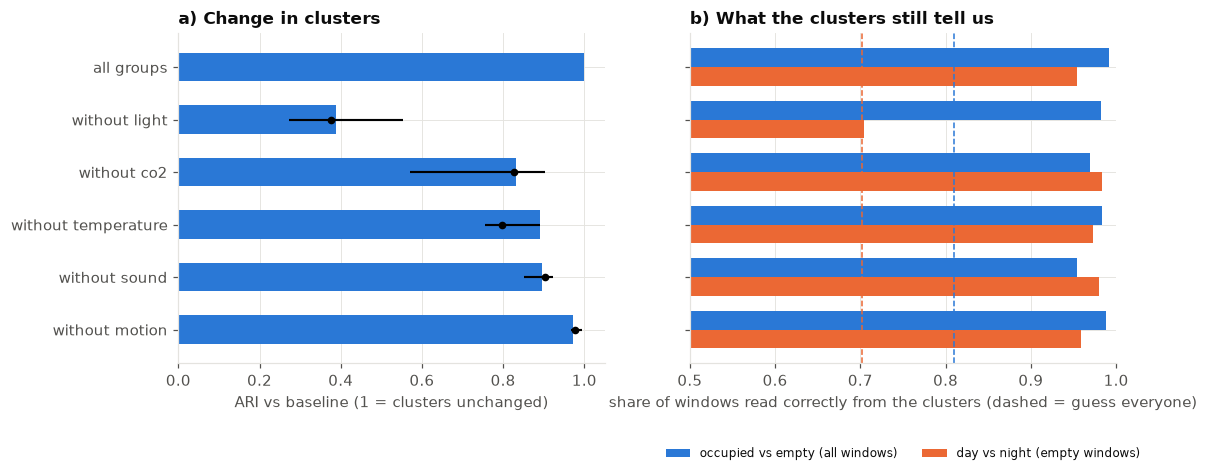

In [38]:
drops = sorted([f"drop {g}" for g in groups], key=lambda n: res.loc[n, "ARI"])  # drop-one variants, most influential first
order = ["all groups"] + drops                                                  # all-groups row on top as the reference
y = np.arange(len(order))                                                       # vertical positions
names = ["all groups"] + [o.replace("drop ", "without ") for o in drops]        # readable row labels
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)                    # sharey: both panels use the same row labels, written once on the left

ax[0].barh(y, res.loc[order, "ARI"], color="#2a78d6", height=0.55)             # bars: ARI vs baseline, all days
sub = res.loc[drops]                                                            # the rows that have a leave-one-day-out range
ax[0].errorbar(sub["ARI_median"], y[1:], xerr=[sub["ARI_median"] - sub["ARI_min"], sub["ARI_max"] - sub["ARI_median"]], fmt="o", color="black", ms=4)   # dot: median over days; line: min to max
ax[0].set_yticks(y); ax[0].set_yticklabels(names); ax[0].invert_yaxis()
ax[0].set_xlim(0, 1.05); ax[0].set_xlabel("ARI vs baseline (1 = clusters unchanged)"); ax[0].set_title("a) Change in clusters", loc="left")

h = 0.36                                                                        # bar thickness in panel b
ax[1].barh(y - h/2, res.loc[order, "occupancy_readout"], height=h, color="#2a78d6", label="occupied vs empty (all windows)")   # occupancy read-out
ax[1].barh(y + h/2, res.loc[order, "daynight_readout"], height=h, color="#eb6834", label="day vs night (empty windows)")      # day/night read-out
ax[1].axvline(guess_occ, color="#2a78d6", ls="--", lw=1)                        # blue dashed: accuracy of guessing "empty" for everyone
ax[1].axvline(guess_day, color="#eb6834", ls="--", lw=1)                        # orange dashed: accuracy of guessing "night" for everyone
ax[1].set_xlim(0.5, 1.0); ax[1].set_xlabel("share of windows read correctly from the clusters (dashed = guess everyone)")
ax[1].set_title("b) What the clusters still tell us", loc="left"); ax[1].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)

Path("figures").mkdir(exist_ok=True)                                            # make the folder if it is missing
fig.savefig("figures/fig_r3_sensor_ablation.png", dpi=300, bbox_inches="tight") # high resolution for the A0 poster
plt.show()

share of all variation shown in this plane: 0.65


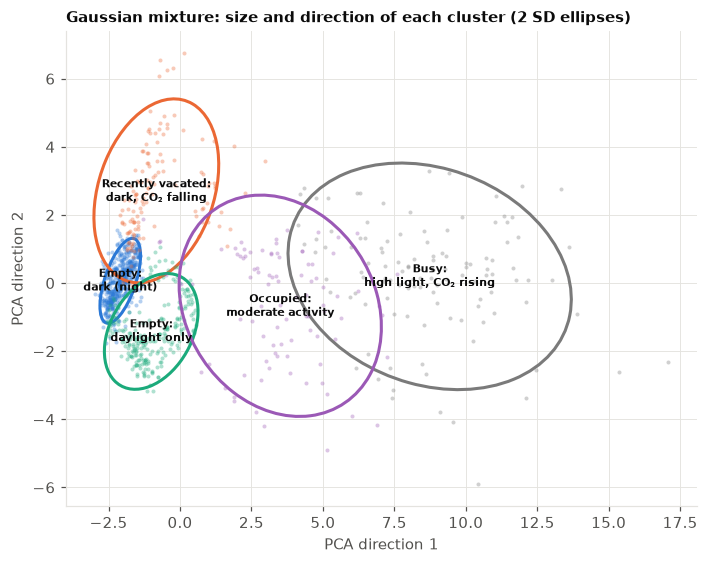

,cluster,windows,axis ratio (plane),angle (deg),main spread in 24-D is mostly,its share
0,"Busy: high light, CO₂ rising",115,1.57,166.81,sound,0.83
1,Empty: dark (night),468,2.50,67.40,temperature,1.00
2,"Recently vacated: dark, CO₂ falling",129,1.44,63.53,light,0.44
3,Empty: daylight only,240,1.43,48.05,temperature,0.77
4,Occupied: moderate activity,92,1.24,147.08,motion,0.43


In [39]:
from matplotlib.patches import Ellipse                                      # draws an ellipse on a plot
from sklearn.decomposition import PCA                                         # finds the directions of largest variation
pca2 = PCA(2).fit(X)                                                          # the 2 directions of largest variation in the 24 scaled features
Z = pca2.transform(X)                                                         # every window as a point in that plane
print("share of all variation shown in this plane:", pca2.explained_variance_ratio_.sum().round(2))

# give each mixture component the name of the Person 2 cluster that most of its windows belong to
comp_name = {k: pd.Series(base_name[lab_gmm == k]).mode()[0] for k in range(K)}     # most common baseline name in each component

rows = []
fig, ax = plt.subplots(figsize=(7.4, 5.6))
colours = ["#7a7a7a", "#2a78d6", "#eb6834", "#1baa7b", "#9b59b6"]
for k in range(K):
    P2 = pca2.components_                                                      # 2 x 24 projection matrix
    S2 = P2 @ gmm.covariances_[k] @ P2.T                                       # the cluster's 24-D covariance seen in the 2-D plane
    m2 = P2 @ (gmm.means_[k] - pca2.mean_)                                     # the cluster's centre in the plane
    w, v = np.linalg.eigh(S2); w, v = w[::-1], v[:, ::-1]                      # eigenvalues (spread) and eigenvectors (directions), longest first
    angle = np.degrees(np.arctan2(v[1, 0], v[0, 0])) % 180                     # direction of the longest axis, 0-180 degrees
    ax.scatter(Z[lab_gmm == k, 0], Z[lab_gmm == k, 1], s=7, alpha=0.35, color=colours[k], linewidths=0)
    ax.add_patch(Ellipse(m2, 4*np.sqrt(w[0]), 4*np.sqrt(w[1]), angle=angle, fill=False, color=colours[k], lw=2))   # 2 standard deviations
    ax.annotate(comp_name[k].replace(": ", ":\n"), m2, ha="center", va="center", fontsize=7, fontweight="bold")
    # direction of the cluster's main spread in the FULL 24-D space: which sensor groups load on it?
    wf, vf = np.linalg.eigh(gmm.covariances_[k]); top = vf[:, -1] ** 2          # squared loadings of the longest axis (sum to 1)
    share = {g: float(sum(top[cols.index(c)] for c in groups[g])) for g in groups}
    rows.append({"cluster": comp_name[k], "windows": int((lab_gmm == k).sum()),
                 "axis ratio (plane)": np.sqrt(w[0] / w[1]), "angle (deg)": angle,
                 "main spread in 24-D is mostly": max(share, key=share.get), "its share": max(share.values())})
ax.set_xlabel("PCA direction 1"); ax.set_ylabel("PCA direction 2")
ax.set_title("Gaussian mixture: size and direction of each cluster (2 SD ellipses)", loc="left", fontsize=10)
fig.savefig("figures/fig_r3_gaussian_direction.png", dpi=300, bbox_inches="tight")
plt.show()
pd.DataFrame(rows).round(2)

**Reading it.**
- **Size matters more than direction.** The ellipses are very different sizes: the night-time cluster is small and tight, while the busy and occupied clusters are huge and spread out. k-means treats every cluster as the same size, so this is the clearest sign that its round, equal-size assumption is only an approximation here.
- **Direction.** Only the night cluster is clearly elongated (axis ratio about 2.5, tilted at about 67 degrees). The others are only mildly stretched (ratios 1.2 to 1.6), so they are closer to round than to long thin ellipses. Directions differ between clusters (angles from about 48 to 167 degrees), so there is no single shared direction of spread.
- **What each cluster stretches along, in the full 24 dimensions** (last two table columns): the busy cluster mostly along sound (83% of that direction), the night cluster along temperature, and the daylight cluster along temperature (77%). For the "recently vacated" and "occupied" clusters the direction is a mixture (light 44%, motion 43%), so do not read much into those two.
- **Overlap.** The occupied and busy ellipses overlap heavily, as do the night and recently-vacated ones. Windows near those boundaries could go either way, which is consistent with the mixture agreeing with k-means at ARI 0.76 rather than near 1.
- **Caveat.** This plane shows 65% of the variation, so ellipses that overlap here may be separated in the other dimensions.


## 3.5 Relationships Between Sensor Groups

Different sensor types may capture related aspects of room conditions. For example, changes in PIR motion, sound and CO₂ measurements may occur during similar periods, while temperature and CO₂ may reflect broader environmental changes.

This investigation examines the relationships between sensor groups to understand whether they provide independent information or capture overlapping patterns.

Ridge Regression and Random Forest models are used to investigate how well one sensor group can be estimated from other sensor measurements. Model performance is assessed using a leave-one-day-out evaluation approach and the coefficient of determination (R²).

Higher predictive performance suggests that the target sensor group shares information with the other measurements. However, this does not establish a causal relationship between the sensors.

Understanding these relationships helps interpret the sensor contribution results and identify possible redundancy within the feature representation.


In [40]:
from sklearn.linear_model import Ridge                                       # straight-line regression with a small penalty (stable when columns are correlated)
from sklearn.ensemble import RandomForestRegressor                           # an ensemble of decision trees, can follow nonlinear patterns
from sklearn.metrics import r2_score                                         # the score: share of variation predicted

day = W["date"].to_numpy()                                                   # the recording day of every window
G = list(groups)                                                             # the five group names

def cv_r2(sources, target, make_model):                                      # predict `target` group from `sources` groups, always on an unseen day
    A = X[sum([groups[g] for g in sources], [])].to_numpy()                  # input columns
    Y = X[groups[target]].to_numpy(); pred = np.zeros_like(Y)                # columns to predict
    for d in sorted(set(day)):                                               # for each day...
        test = day == d                                                      # ...that day is the test set
        pred[test] = make_model().fit(A[~test], Y[~test]).predict(A[test])   # ...train on all other days, predict this one
    return r2_score(Y, pred, multioutput="uniform_average")                  # average R2 across the target's columns

ridge = lambda: Ridge(alpha=1.0)
forest = lambda: RandomForestRegressor(200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)

pair = pd.DataFrame({t: {s: cv_r2([s], t, ridge) if s != t else np.nan for s in G} for t in G})    # rows = source, columns = target
rest = pd.DataFrame({"straight-line (ridge)": {t: cv_r2([g for g in G if g != t], t, ridge) for t in G},
                     "random forest":        {t: cv_r2([g for g in G if g != t], t, forest) for t in G}})   # all other groups -> target
print("(a) R2 predicting the column group from the row group, on unseen days:"); print(pair.round(2).to_string())
print("\n(b) R2 predicting each group from ALL the other groups, on unseen days:"); print(rest.round(2).to_string())

(a) R2 predicting the column group from the row group, on unseen days:
             temperature  light  sound   co2  motion
temperature          NaN   0.28   0.30  0.28    0.38
light               0.18    NaN   0.60  0.35    0.49
sound               0.14   0.39    NaN  0.34    0.58
co2                 0.29   0.29   0.51   NaN    0.49
motion              0.12   0.35   0.55  0.27     NaN

(b) R2 predicting each group from ALL the other groups, on unseen days:
             straight-line (ridge)  random forest
temperature                   0.26           0.24
light                         0.13           0.48
sound                         0.58           0.66
co2                           0.45           0.39
motion                        0.57           0.60


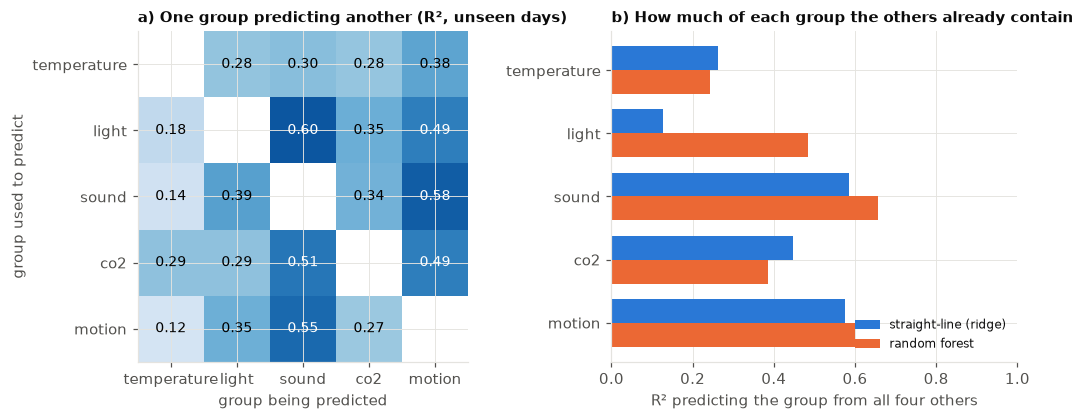

,R2 from the others (forest),ARI when dropped
temperature,0.24,0.89
light,0.48,0.39
sound,0.66,0.89
co2,0.39,0.83
motion,0.60,0.97


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.1, 1]})
im = ax[0].imshow(pair.to_numpy(float), cmap="Blues", vmin=0, vmax=0.7)       # colour = R2 (negative values shown as the lightest colour)
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(G); ax[0].set_yticks(range(5)); ax[0].set_yticklabels(G)
for i in range(5):
    for j in range(5):
        if i != j: ax[0].text(j, i, f"{pair.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if pair.iloc[i, j] > 0.4 else "black")
ax[0].set_xlabel("group being predicted"); ax[0].set_ylabel("group used to predict")
ax[0].set_title("a) One group predicting another (R², unseen days)", loc="left", fontsize=10)
y = np.arange(5); h = 0.38
ax[1].barh(y - h/2, rest["straight-line (ridge)"], h, color="#2a78d6", label="straight-line (ridge)")
ax[1].barh(y + h/2, rest["random forest"], h, color="#eb6834", label="random forest")
ax[1].set_yticks(y); ax[1].set_yticklabels(G); ax[1].invert_yaxis(); ax[1].set_xlim(0, 1)
ax[1].set_xlabel("R² predicting the group from all four others"); ax[1].legend(frameon=False, fontsize=8, loc="lower right")
ax[1].set_title("b) How much of each group the others already contain", loc="left", fontsize=10)
fig.savefig("figures/fig_r3_group_dependence.png", dpi=300, bbox_inches="tight")
pair.round(4).to_csv("dependence_pairwise.csv"); rest.round(4).to_csv("dependence_all_others.csv")   # saved for Person 6
plt.show()
cmp = pd.DataFrame({"R2 from the others (forest)": rest["random forest"], "ARI when dropped": [res.loc[f"drop {g}", "ARI"] for g in G]}, index=G)
cmp.round(2)

**Reading it.**
- **Sound and motion are the most redundant.** Each can be predicted from the other groups with R² of about 0.6 (sound 0.58 to 0.66, motion 0.57 to 0.60). The strongest single pairs are light to sound (0.60) and sound to motion (0.58), and motion to sound (0.55). This fits the ablation: removing motion changed the clusters least (ARI 0.97), because the other groups largely stand in for it.
- **Temperature is the least predictable** (R² about 0.25), so it carries information the others do not. But removing it barely changes the clusters (ARI 0.89), so unique information is not the same as important information for these clusters.
- **Light depends on the others in a curved way.** A straight-line model predicts light poorly (0.13) but the random forest does much better (0.48), so the relationship is nonlinear, plausibly because daylight switches light on and off. Light is still the group whose removal changes the clusters most (ARI 0.39).
- **CO₂** sits in the middle (0.39 to 0.45).
- **Limits.** Prediction is not causation: two groups can predict each other because the same thing (the time of day, or someone being in the room) drives both. Sound and motion in particular both respond to people. With five groups there is no clean rule linking redundancy to influence, so describe it as "consistent with" and not as an explanation.


## 3.6 Summary of Validation and Sensor Contribution

This section evaluates the reliability of the discovered clustering structure and examines how it is influenced by the clustering method, feature representation and sensor measurements.

The stability analysis assesses whether similar patterns are identified under different initialisation and recording-period conditions. The method and representation comparisons investigate whether the discovered structure is dependent on particular analytical choices.

Finally, sensor ablation and sensor-group relationship analysis provide insight into the contribution and potential overlap of different sensor measurements.

Together, these investigations provide a stronger basis for interpreting the five-cluster solution and identifying which sensor groups are most informative for distinguishing recurring room conditions.


In [42]:
# MERGE FIX: Section 3 reloaded W from windows_5min.csv (text 'start', no cluster columns).
# Section 4 was written for the Section 1-2 table, so restore it.
W = W_main.copy()
assert len(W) == len(X_node) == len(W_lab), 'W, X_node and W_lab must describe the same windows'
assert pd.api.types.is_datetime64_any_dtype(W['start'])
print('Section 4 table restored:', W.shape)


Section 4 table restored: (1044, 39)



# 4. Anomaly Detection

## 4.1 Objective and Research Question

Following the identification of recurring room-usage patterns through clustering, this section investigates unusual sensor behaviour within those patterns.

The main research question is:

**Which five-minute observation windows exhibit unusual sensor behaviour relative to their identified room-usage patterns, and can these observations be distinguished as potential unusual room behaviour, sensor faults or data-quality issues?**

An observation is considered potentially anomalous when its sensor measurements differ substantially from the typical behaviour of its assigned cluster.

This distinction is important because a globally unusual observation may simply represent a legitimate room state. For example, a busy room may appear unusual when compared with predominantly empty-room observations.

Therefore, the analysis considers both global anomaly detection and state-aware anomaly detection. The K-Means clusters identified in Section 2 provide the reference room states.

Occupancy labels are excluded from anomaly detection and are used only for subsequent evaluation and interpretation.



### 4.2 Anomaly Detection Methods

Four anomaly scores are investigated:

1. **Global Isolation Forest:** Provides a baseline by identifying observations that are unusual across the complete dataset.
2. **Local Outlier Factor (LOF):** Measures how locally isolated an observation is compared with other observations belonging to the same cluster.
3. **Distance to Cluster Centroid:** Measures how far an observation is from the centre of its assigned cluster, scaled by the median distance within that cluster.
4. **Within-Cluster Isolation Forest:** Fits a separate Isolation Forest model for each cluster to identify unusual observations relative to their own room state.

The node-level sensor representation is used initially because it retains individual sensor information.

Since the four scores have different numerical scales, they are converted into percentile ranks. The three state-aware methods are then combined using a consensus rule: an observation is flagged when at least two of the three state-aware scores fall within their respective top 5%.

The 5% threshold is an exploratory choice rather than a known proportion of true anomalies. Its sensitivity is examined later in this section.


In [43]:

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import KMeans

# Recreate the same K-Means assignments used in Section 2
XA = X_node.values

km_anomaly = KMeans(
    n_clusters=K_FINAL,
    n_init=20,
    random_state=RANDOM_SEED
)

cluster_labels = km_anomaly.fit_predict(XA)

# Store assignments in W for subsequent analysis
W["cluster"] = cluster_labels
W["cluster_name"] = W["cluster"].map(CLUSTER_NAMES)

STATE_SCORES = ["lof", "centroid", "iso_state"]

def anomaly_scores(X, clusters, lof_k=20, seed=42):

    X = np.asarray(X)
    clusters = np.asarray(clusters)

    scores = pd.DataFrame(index=W.index)

    # 1. Global Isolation Forest
    global_if = IsolationForest(
        n_estimators=500,
        random_state=seed
    )
    global_if.fit(X)
    scores["iso_global"] = -global_if.score_samples(X)

    # 2. State-aware Local Outlier Factor
    scores["lof"] = np.nan

    for c in np.unique(clusters):
        mask = clusters == c
        n = mask.sum()

        if n < 3:
            raise ValueError(
                f"Cluster {c} has too few observations for LOF."
            )

        k = min(lof_k, n - 1)

        lof = LocalOutlierFactor(n_neighbors=k)
        scores.loc[mask, "lof"] = (
            -lof.fit(X[mask]).negative_outlier_factor_
        )

    # 3. Distance to own cluster centroid
    centres = {
        c: X[clusters == c].mean(axis=0)
        for c in np.unique(clusters)
    }

    distances = np.array([
        np.linalg.norm(X[i] - centres[clusters[i]])
        for i in range(len(X))
    ])

    distance_series = pd.Series(distances, index=W.index)

    median_distances = distance_series.groupby(
        clusters
    ).transform("median").clip(lower=1e-9)

    scores["centroid"] = distance_series / median_distances

    # 4. Within-cluster Isolation Forest
    scores["iso_state"] = np.nan

    for c in np.unique(clusters):
        mask = clusters == c

        state_if = IsolationForest(
            n_estimators=500,
            random_state=seed
        )
        state_if.fit(X[mask])

        scores.loc[mask, "iso_state"] = (
            -state_if.score_samples(X[mask])
        )

    return scores


# Calculate anomaly scores
A = anomaly_scores(
    XA,
    cluster_labels,
    lof_k=20
)

# Global Isolation Forest: rank across the complete dataset
A_pct = pd.DataFrame(index=A.index)

A_pct["iso_global"] = A["iso_global"].rank(pct=True)

# State-aware scores: rank within each assigned cluster
for score in STATE_SCORES:
    A_pct[score] = A[score].groupby(
        W["cluster"]
    ).rank(pct=True)

print("Cluster sizes:")
print(W["cluster"].value_counts().sort_index())

print("\nAnomaly scores:")
display(A.head())

print("\nSpearman correlation:")
display(A.corr(method="spearman").round(2))


Cluster sizes:
cluster
0     82
1    545
2     88
3    216
4    113
Name: count, dtype: int64

Anomaly scores:


,iso_global,lof,centroid,iso_state
0,0.594830,1.201911,1.455836,0.548477
1,0.571997,1.113310,1.308560,0.517223
2,0.536271,2.199407,2.111352,0.701155
3,0.497425,1.979840,1.227358,0.652661
4,0.526358,1.955540,1.958049,0.691934



Spearman correlation:


,iso_global,lof,centroid,iso_state
iso_global,1.00,0.20,0.42,0.73
lof,0.20,1.00,0.57,0.50
centroid,0.42,0.57,1.00,0.66
iso_state,0.73,0.50,0.66,1.00



### 4.3 Global versus State-Aware Anomaly Detection

Global anomaly detection provides a useful baseline, but it may identify legitimate room states as unusual because different room-usage patterns have different sensor characteristics.

To investigate this limitation, the global Isolation Forest results are compared with the state-aware consensus.

Each detector uses a top 5% threshold based on its anomaly score. For the state-aware approach, a window is flagged when at least two of the three detectors agree.

The comparison examines how anomaly flags are distributed across the five discovered room-usage clusters.


In [44]:

TOP = 0.05

# Count how many state-aware detectors flag each window
votes = (
    A_pct[STATE_SCORES] >= 1 - TOP
).sum(axis=1)

# Consensus: at least two out of three detectors agree
W["anomaly"] = votes >= 2
W["anomaly_votes"] = votes

# Global Isolation Forest baseline
global_flags = A_pct["iso_global"] >= 1 - TOP

# Compare anomaly rates across room-usage clusters
cluster_order = list(
    W["cluster_name"].drop_duplicates()
)

comparison = pd.DataFrame({
    "Global Isolation Forest (%)":
        global_flags.groupby(W["cluster_name"]).mean() * 100,

    "State-aware consensus (%)":
        W["anomaly"].groupby(W["cluster_name"]).mean() * 100
}).reindex(cluster_order)

print(
    f"Global Isolation Forest flagged "
    f"{global_flags.sum()} windows."
)

print(
    f"State-aware consensus flagged "
    f"{W['anomaly'].sum()} windows "
    f"out of {len(W)}."
)

display(comparison.round(2))


Global Isolation Forest flagged 53 windows.
State-aware consensus flagged 35 windows out of 1044.


,Global Isolation Forest (%),State-aware consensus (%)
cluster_name,,
Occupied: moderate activity,9.73,5.31
Empty: daylight only,0.00,4.17
"Busy: high light, CO₂ rising",51.22,6.10
"Recently vacated: dark, CO₂ falling",0.00,1.14
Empty: dark (night),0.00,2.57



### Interpretation

The global Isolation Forest identified 53 potentially unusual windows (5.08% of the dataset), whereas the state-aware consensus identified 36 windows (3.45%). This difference suggests that the choice of reference population influences which observations are considered unusual.

The cluster-level comparison provides further insight. The global method flagged 51.22% of observations in the busy, high-light and rising-CO₂ cluster, while it did not flag observations in the two empty-room clusters or the recently vacated cluster. This suggests that the global model may be particularly sensitive to environmental differences between room-usage patterns.

In contrast, the state-aware consensus identified potentially unusual observations across all five clusters. This indicates that unusual behaviour can occur within different room states rather than being limited to one globally distinctive pattern.

The relatively low correlation between global Isolation Forest and LOF (Spearman correlation = 0.20) further demonstrates that different detection methods capture different aspects of unusual behaviour.

Overall, the results support using state-aware detection alongside a global baseline. However, flagged observations represent candidates for further investigation rather than confirmed anomalies or sensor faults.


### 4.4 Sensor Deviations and Potential Data-Quality Issues

To investigate which sensor features contributed to the flagged observations, robust deviations were calculated relative to the median feature values within each cluster. This provides a comparison against the typical behaviour of the corresponding room-usage pattern, rather than against the entire dataset.

The state-aware consensus identified 36 potentially unusual windows. Among these, `S1_Sound_mean` and `S4_Temp_mean` were the strongest individual feature deviations in five windows each, followed by `S3_Sound_mean` in four windows. Other contributing features included light measurements, CO₂ levels and sound measurements from different sensor locations. This indicates that unusual observations were associated with different aspects of the room environment rather than one consistently dominant sensor.

The number of features with a robust deviation of at least three varied across flagged windows. Twelve windows had no individual feature exceeding this threshold, while some observations showed deviations across several features. Therefore, an observation can be flagged by the anomaly-detection methods without having one feature that independently exceeds the sensor-deviation threshold.

These results help identify which measurements may warrant further inspection. However, a large deviation does not confirm a sensor fault. It may reflect genuine environmental variation, unusual room activity, measurement noise or a data-quality issue. The analysis therefore treats these observations as candidates for investigation rather than confirmed sensor failures.

In [45]:
print(W.columns.tolist())

['segment', 'win', 'start', 'n_readings', 'S1_Temp_mean', 'S1_Temp_delta', 'S2_Temp_mean', 'S2_Temp_delta', 'S3_Temp_mean', 'S3_Temp_delta', 'S4_Temp_mean', 'S4_Temp_delta', 'S1_Light_mean', 'S2_Light_mean', 'S3_Light_mean', 'S4_Light_mean', 'S1_Sound_mean', 'S1_Sound_max', 'S2_Sound_mean', 'S2_Sound_max', 'S3_Sound_mean', 'S3_Sound_max', 'S4_Sound_mean', 'S4_Sound_max', 'CO2_excess_mean', 'CO2_slope_mean', 'S6_PIR_frac', 'S7_PIR_frac', 'temp_mean', 'temp_delta', 'light_mean', 'sound_mean', 'sound_max', 'pir_frac', 'date', 'hour', 'cluster', 'dist_to_centroid', 'cluster_name', 'anomaly', 'anomaly_votes']


In [46]:

# Identify sensor features for anomaly interpretation

sensor_features = [
    col for col in X_node.columns
]

# Calculate robust cluster-specific deviations
# using median and median absolute deviation (MAD)

sensor_deviations = pd.DataFrame(
    index=W.index,
    columns=sensor_features,
    dtype=float
)

for cluster_id in W["cluster"].unique():

    mask = W["cluster"] == cluster_id

    cluster_data = X_node.loc[mask, sensor_features]

    median = cluster_data.median()
    mad = (cluster_data - median).abs().median()

    # Avoid division by zero for constant features
    mad = mad.replace(0, np.nan)

    deviations = (
        X_node.loc[mask, sensor_features] - median
    ).abs() / (1.4826 * mad)

    sensor_deviations.loc[mask] = deviations

sensor_deviations = sensor_deviations.fillna(0)

# Identify the strongest sensor driver for each window
W["strongest_sensor"] = (
    sensor_deviations.idxmax(axis=1)
)

W["max_sensor_deviation"] = (
    sensor_deviations.max(axis=1)
)

print("Sensor deviation summary:")
display(
    sensor_deviations.describe().round(2)
)

print("\nStrongest sensor drivers among flagged windows:")

display(
    W.loc[
        W["anomaly"],
        "strongest_sensor"
    ].value_counts().to_frame("Flagged windows")
)


Sensor deviation summary:


,S1_Temp_mean,S2_Temp_mean,S3_Temp_mean,S4_Temp_mean,S1_Temp_delta,S2_Temp_delta,S3_Temp_delta,S4_Temp_delta,S1_Light_mean,S2_Light_mean,...,S3_Sound_mean,S4_Sound_mean,S1_Sound_max,S2_Sound_max,S3_Sound_max,S4_Sound_max,CO2_excess_mean,CO2_slope_mean,S6_PIR_frac,S7_PIR_frac
count,1044.00,1044.00,1044.00,1044.00,1044.0,1044.00,1044.00,1044.00,1044.00,1044.00,...,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00
mean,0.80,0.83,0.80,0.80,0.0,0.15,0.03,0.14,0.50,0.84,...,1.15,0.98,0.26,0.78,0.42,0.70,1.07,0.27,0.13,0.21
std,0.74,0.79,0.67,0.65,0.0,0.80,0.15,0.33,1.42,3.54,...,1.89,1.24,1.41,1.72,1.22,0.79,3.23,0.69,0.35,0.67
min,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.35,0.34,0.30,0.34,0.0,0.00,0.00,0.00,0.00,0.00,...,0.34,0.32,0.00,0.00,0.00,0.17,0.00,0.00,0.00,0.00
50%,0.67,0.67,0.67,0.67,0.0,0.00,0.00,0.00,0.00,0.00,...,0.67,0.67,0.00,0.67,0.00,0.67,0.37,0.00,0.00,0.00
75%,1.01,1.01,1.09,1.17,0.0,0.00,0.00,0.00,0.41,0.37,...,1.35,1.03,0.00,0.68,0.40,0.69,0.71,0.09,0.00,0.00
max,8.96,6.23,4.63,6.02,0.0,14.05,1.35,2.14,11.20,25.62,...,29.42,9.25,31.02,20.30,16.31,7.72,36.80,6.25,2.28,5.40



Strongest sensor drivers among flagged windows:


,Flagged windows
strongest_sensor,
S1_Sound_mean,5
S4_Temp_mean,5
CO2_excess_mean,3
S1_Temp_mean,2
S3_Light_mean,2
S2_Temp_mean,2
S4_Light_mean,2
S3_Sound_mean,2
S4_Sound_mean,2


In [47]:

# Summarise sensor drivers for flagged windows

flagged_windows = W.loc[W["anomaly"]].copy()

flagged_windows["sensor_groups_affected"] = (
    sensor_deviations.loc[W["anomaly"]]
    .ge(3)
    .sum(axis=1)
)

print("Number of flagged windows:", len(flagged_windows))

print("\nSensor groups affected:")

display(
    flagged_windows[
        "sensor_groups_affected"
    ].value_counts().sort_index().to_frame("Windows")
)

print("\nExamples of flagged observations:")

display(
    flagged_windows[
        [
            "start",
            "cluster_name",
            "anomaly_votes",
            "strongest_sensor",
            "max_sensor_deviation",
            "sensor_groups_affected"
        ]
    ].head(10)
)


Number of flagged windows: 35

Sensor groups affected:


,Windows
sensor_groups_affected,
0,13
1,6
2,1
3,1
4,3
5,1
6,7
7,3



Examples of flagged observations:


,start,cluster_name,anomaly_votes,strongest_sensor,max_sensor_deviation,sensor_groups_affected
0,2017-12-22 10:49:41,Occupied: moderate activity,2,S1_Temp_mean,3.649237,2
2,2017-12-22 10:59:54,Empty: daylight only,3,S1_Sound_mean,124.346607,7
3,2017-12-22 11:05:00,Empty: daylight only,2,S1_Sound_mean,36.708479,6
4,2017-12-22 11:10:06,Empty: daylight only,3,S1_Sound_mean,122.781809,6
5,2017-12-22 11:14:42,Empty: daylight only,2,S1_Sound_mean,83.176935,6
6,2017-12-22 11:19:49,Empty: daylight only,3,S1_Sound_mean,126.126301,6
7,2017-12-22 11:24:55,Occupied: moderate activity,2,S7_PIR_frac,2.697963,0
12,2017-12-22 11:55:02,"Busy: high light, CO₂ rising",3,S3_Light_mean,20.284827,7
13,2017-12-22 12:00:09,Occupied: moderate activity,2,S2_Temp_mean,2.357785,0
15,2017-12-22 12:09:51,Occupied: moderate activity,2,S2_Temp_mean,2.614092,0


In [48]:
flagged_windows = W.loc[W["anomaly"]].copy()

flagged_windows["features_affected"] = (
    sensor_deviations.loc[W["anomaly"]].ge(3).sum(axis=1)
)

display(
    flagged_windows[
        [
            "start",
            "cluster_name",
            "anomaly_votes",
            "strongest_sensor",
            "max_sensor_deviation",
            "features_affected"
        ]
    ].head(10)
)

,start,cluster_name,anomaly_votes,strongest_sensor,max_sensor_deviation,features_affected
0,2017-12-22 10:49:41,Occupied: moderate activity,2,S1_Temp_mean,3.649237,2
2,2017-12-22 10:59:54,Empty: daylight only,3,S1_Sound_mean,124.346607,7
3,2017-12-22 11:05:00,Empty: daylight only,2,S1_Sound_mean,36.708479,6
4,2017-12-22 11:10:06,Empty: daylight only,3,S1_Sound_mean,122.781809,6
5,2017-12-22 11:14:42,Empty: daylight only,2,S1_Sound_mean,83.176935,6
6,2017-12-22 11:19:49,Empty: daylight only,3,S1_Sound_mean,126.126301,6
7,2017-12-22 11:24:55,Occupied: moderate activity,2,S7_PIR_frac,2.697963,0
12,2017-12-22 11:55:02,"Busy: high light, CO₂ rising",3,S3_Light_mean,20.284827,7
13,2017-12-22 12:00:09,Occupied: moderate activity,2,S2_Temp_mean,2.357785,0
15,2017-12-22 12:09:51,Occupied: moderate activity,2,S2_Temp_mean,2.614092,0


### 4.5 Evaluation Against Occupancy Labels

The detected anomalies are compared with the recorded occupancy labels to investigate whether unusual sensor behaviour is associated with occupied periods, empty periods or occupancy transitions.

The analysis compares anomaly rates across empty and occupied windows and examines whether flagged observations occur more frequently during windows containing occupancy transitions.

Occupancy labels are used exclusively for evaluation and interpretation, not as inputs to the anomaly-detection models.

In [49]:

# Evaluate detected anomalies against occupancy labels

# Confirm that feature windows and label windows are aligned
assert len(W) == len(L), "Window and label counts do not match."

evaluation = W[
    ["start", "cluster_name", "anomaly", "anomaly_votes"]
].copy()

# Add separately stored occupancy labels for evaluation only
evaluation["occupied"] = L["occupied"].astype(bool).to_numpy()
evaluation["occ_mode"] = L["occ_mode"].to_numpy()
evaluation["transition"] = L["transition"].astype(bool).to_numpy()

# 1. Compare anomaly rates in empty and occupied windows
print("Anomaly detection by occupancy status:")

occupancy_summary = (
    evaluation.groupby("occupied")["anomaly"]
    .agg(
        windows="count",
        flagged="sum",
        anomaly_rate="mean"
    )
)

occupancy_summary["anomaly_rate"] *= 100

display(occupancy_summary.round(2))

# 2. Compare anomaly rates during transition and non-transition windows
print("\nAnomaly detection by occupancy transition:")

transition_summary = (
    evaluation.groupby("transition")["anomaly"]
    .agg(
        windows="count",
        flagged="sum",
        anomaly_rate="mean"
    )
)

transition_summary["anomaly_rate"] *= 100

display(transition_summary.round(2))

# 3. Compare recorded head-counts in flagged and non-flagged windows
print("\nRecorded occupancy counts by anomaly status:")

headcount_summary = pd.crosstab(
    evaluation["anomaly"],
    evaluation["occ_mode"],
    rownames=["Anomaly flagged"],
    colnames=["Recorded occupants"]
)

display(headcount_summary)

# 4. Inspect flagged observations
print("\nExamples of flagged observations and their occupancy labels:")

display(
    evaluation.loc[
        evaluation["anomaly"],
        [
            "start",
            "cluster_name",
            "anomaly_votes",
            "occupied",
            "occ_mode",
            "transition"
        ]
    ].head(10)
)


Anomaly detection by occupancy status:


,windows,flagged,anomaly_rate
occupied,,,
False,846,18,2.13
True,198,17,8.59



Anomaly detection by occupancy transition:


,windows,flagged,anomaly_rate
transition,,,
False,1024,33,3.22
True,20,2,10.00



Recorded occupancy counts by anomaly status:


Recorded occupants,0,1,2,3
Anomaly flagged,,,,
False,832,40,70,67
True,18,8,4,5



Examples of flagged observations and their occupancy labels:


,start,cluster_name,anomaly_votes,occupied,occ_mode,transition
0,2017-12-22 10:49:41,Occupied: moderate activity,2,True,1,False
2,2017-12-22 10:59:54,Empty: daylight only,3,True,1,False
3,2017-12-22 11:05:00,Empty: daylight only,2,True,1,False
4,2017-12-22 11:10:06,Empty: daylight only,3,True,1,False
5,2017-12-22 11:14:42,Empty: daylight only,2,True,1,False
6,2017-12-22 11:19:49,Empty: daylight only,3,True,1,False
7,2017-12-22 11:24:55,Occupied: moderate activity,2,True,1,True
12,2017-12-22 11:55:02,"Busy: high light, CO₂ rising",3,True,2,False
13,2017-12-22 12:00:09,Occupied: moderate activity,2,True,2,False
15,2017-12-22 12:09:51,Occupied: moderate activity,2,True,2,False


In [50]:

# Check anomaly counts and occupancy-label alignment

print("Total windows:", len(W))
print("Flagged in W:", W["anomaly"].sum())
print("Flagged in evaluation:", evaluation["anomaly"].sum())

print("\nMissing occupancy labels:")
print(evaluation["occupied"].isna().sum())

print("\nAnomaly and occupancy counts:")
display(
    pd.crosstab(
        evaluation["anomaly"],
        evaluation["occupied"],
        dropna=False
    )
)


Total windows: 1044
Flagged in W: 35
Flagged in evaluation: 35

Missing occupancy labels:
0

Anomaly and occupancy counts:


occupied,False,True
anomaly,,
False,828,181
True,18,17


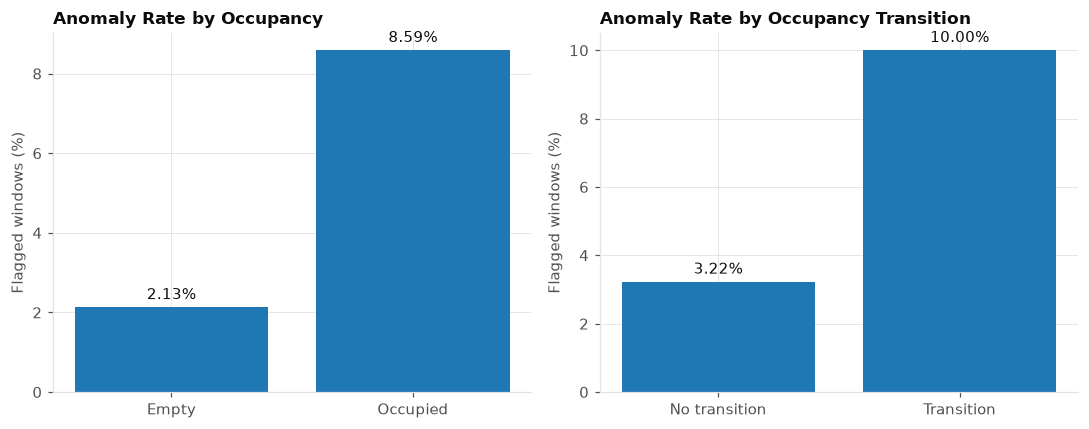

In [51]:

# Visualise anomaly rates against occupancy labels

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Occupancy comparison
occ_rates = (
    evaluation.groupby("occupied")["anomaly"].mean() * 100
)

axes[0].bar(
    ["Empty", "Occupied"],
    [occ_rates.get(False, 0), occ_rates.get(True, 0)]
)

axes[0].set_title("Anomaly Rate by Occupancy")
axes[0].set_ylabel("Flagged windows (%)")

# Transition comparison
trans_rates = (
    evaluation.groupby("transition")["anomaly"].mean() * 100
)

axes[1].bar(
    ["No transition", "Transition"],
    [trans_rates.get(False, 0), trans_rates.get(True, 0)]
)

axes[1].set_title("Anomaly Rate by Occupancy Transition")
axes[1].set_ylabel("Flagged windows (%)")

for ax in axes:
    ax.bar_label(
        ax.containers[0],
        fmt="%.2f%%",
        padding=3
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


Global IF flags 53 windows; 79% of them are in the 'Busy' cluster. Consensus flags 35 windows.


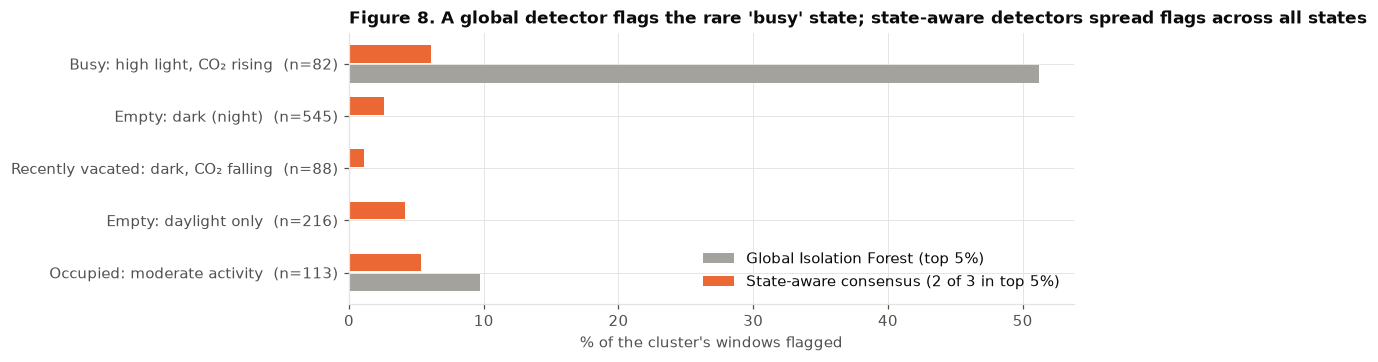

,Global Isolation Forest,State-aware consensus
cluster_name,,
"Busy: high light, CO₂ rising",51.2,6.1
Empty: dark (night),0.0,2.6
"Recently vacated: dark, CO₂ falling",0.0,1.1
Empty: daylight only,0.0,4.2
Occupied: moderate activity,9.7,5.3


In [52]:
TOP = 0.05
votes = (A_pct[STATE_SCORES] >= 1 - TOP).sum(axis=1)
W["anomaly"] = votes >= 2          # at least 2 of 3 state-aware detectors
W["anomaly_votes"] = votes
glob = A_pct["iso_global"] >= 1 - TOP

share = pd.DataFrame({"Global Isolation Forest": glob.groupby(W["cluster_name"]).mean() * 100,
                      "State-aware consensus": W["anomaly"].groupby(W["cluster_name"]).mean() * 100}).loc[ORDER]
print(f"Global IF flags {glob.sum()} windows; {100 * W.loc[glob, 'cluster_name'].str.startswith('Busy').mean():.0f}% "
      f"of them are in the 'Busy' cluster. Consensus flags {W['anomaly'].sum()} windows.")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
yy = np.arange(len(ORDER)); h = 0.38
ax.barh(yy + h/2, share.iloc[:, 0], height=h - 0.04, color=C_GREY, label="Global Isolation Forest (top 5%)")
ax.barh(yy - h/2, share.iloc[:, 1], height=h - 0.04, color=C_ORANGE, label="State-aware consensus (2 of 3 in top 5%)")
ax.set_yticks(yy); ax.set_yticklabels([f"{n}  (n={counts[n]})" for n in ORDER]); ax.invert_yaxis()
ax.set_xlabel("% of the cluster's windows flagged"); ax.legend(loc="lower right")
ax.set_title("Figure 8. A global detector flags the rare 'busy' state; state-aware detectors spread flags across all states")
fig.savefig(f"{FIG_DIR}/fig8_global_vs_state.png"); plt.show()
share.round(1)

In [53]:

# Create 30-second sensor quality and evaluation flags
# These flags are used for categorisation and evaluation only.

gap = df["ts"].diff().dt.total_seconds()

flags = pd.DataFrame(index=df.index)

# Identify readings immediately following a gap longer than 65 seconds
flags["after_gap"] = gap.fillna(0) > 65

# Identify PIR activity when the recorded occupancy label is empty.
# This is for evaluation only, not for anomaly detection.
flags["EVAL_pir_when_empty"] = (
    (df[LABEL] == 0) &
    (df[PIR].max(axis=1) == 1)
)

print("Quality flags created successfully:")
display(flags.sum().to_frame("count"))


Quality flags created successfully:


,count
after_gap,8
EVAL_pir_when_empty,24


In [54]:
FAMILY = {c: g for g, cs in FEATURE_GROUPS.items() for c in cs}
NODE = lambda c: c.split("_")[0] if c.startswith("S") else "S5"   # CO2 features are on S5
TEMP_STEP = 0.07   # 1/16 °C after rounding

# robust z-score against own cluster
med = X_node.groupby(W["cluster"]).transform("median")
mad = (X_node - med).abs().groupby(W["cluster"]).transform("median") * 1.4826
Zst = (X_node - med) / mad.clip(lower=0.1)

# 30 s quality flags -> window level
seg_start = df.groupby("segment")["ts"].transform("min")
win_of_row = ((df["ts"] - seg_start).dt.total_seconds() // (WINDOW_MIN * 60)).astype(int)
FW = flags.groupby([df["segment"], win_of_row]).any()
FW.index.names = ["segment", "win"]
Wflags = W[["segment", "win"]].join(FW, on=["segment", "win"]).drop(columns=["segment", "win"]).fillna(False)

def categorise(i, z_thr=3.0, corr_thr=1.5):
    z = Zst.loc[i]
    # drivers, ignoring one-step temperature changes
    drv = [c for c in z.index[z.abs() > z_thr]
           if not (c.endswith("_Temp_delta") and abs(W.at[i, c]) <= TEMP_STEP + 1e-9)]
    if Wflags.at[i, "after_gap"]:
        cat = "Data gap"
    elif not drv:
        cat = "Resolution artefact"
    elif len({FAMILY[c] for c in drv}) >= 2:
        cat = "Multi-sensor behaviour"
    elif len({NODE(c) for c in drv}) >= 2:
        cat = "Room-wide single type"
    elif FAMILY[drv[0]] == "co2":
        cat = "CO₂ only"
    else:
        # one node: do the other sensors on the same desk agree?
        node = NODE(drv[0])
        others = [c for c in z.index if NODE(c) == node and FAMILY[c] != FAMILY[drv[0]]]
        cat = "One node, corroborated" if (z[others].abs() > corr_thr).any() else "One node, isolated"
    drv = sorted(drv, key=lambda c: -abs(z[c]))
    return cat, ", ".join(drv[:4]), len({FAMILY[c] for c in drv})

CATS = ["Multi-sensor behaviour", "Room-wide single type", "One node, corroborated",
        "One node, isolated", "CO₂ only", "Resolution artefact", "Data gap"]
flagged = W.index[W["anomaly"]]
res = pd.DataFrame([categorise(i) for i in flagged], index=flagged,
                   columns=["category", "drivers", "n_sensor_types"])
W["anomaly_category"] = res["category"].reindex(W.index)
W["anomaly_drivers"] = res["drivers"].reindex(W.index)
print(res["category"].value_counts().reindex(CATS, fill_value=0).to_frame("windows"))
res.join(W[["start", "cluster_name"]]).sort_values("start")

                        windows
category                       
Multi-sensor behaviour       14
Room-wide single type         7
One node, corroborated        4
One node, isolated            5
CO₂ only                      2
Resolution artefact           2
Data gap                      1


,category,drivers,n_sensor_types,start,cluster_name
0,Room-wide single type,"S1_Temp_mean, S4_Temp_mean",1,2017-12-22 10:49:41,Occupied: moderate activity
2,Multi-sensor behaviour,"S1_Sound_max, S6_PIR_frac, S1_Sound_mean, S2_S...",3,2017-12-22 10:59:54,Empty: daylight only
3,Multi-sensor behaviour,"S1_Sound_max, CO2_slope_mean, S1_Sound_mean, S...",4,2017-12-22 11:05:00,Empty: daylight only
4,Multi-sensor behaviour,"S1_Sound_max, S1_Sound_mean, CO2_slope_mean, S...",4,2017-12-22 11:10:06,Empty: daylight only
5,Multi-sensor behaviour,"S1_Sound_max, S1_Sound_mean, S6_PIR_frac, CO2_...",4,2017-12-22 11:14:42,Empty: daylight only
6,Multi-sensor behaviour,"S1_Sound_mean, S1_Sound_max, S6_PIR_frac, CO2_...",4,2017-12-22 11:19:49,Empty: daylight only
7,"One node, isolated",S2_Temp_delta,1,2017-12-22 11:24:55,Occupied: moderate activity
12,Multi-sensor behaviour,"S2_Temp_delta, S4_Light_mean, S1_Temp_mean, S4...",3,2017-12-22 11:55:02,"Busy: high light, CO₂ rising"
13,"One node, corroborated",S2_Temp_delta,1,2017-12-22 12:00:09,Occupied: moderate activity
15,"One node, corroborated",S2_Temp_delta,1,2017-12-22 12:09:51,Occupied: moderate activity


##### Check against labels (evaluation only)
If the sorting makes sense, behaviour windows should line up with occupancy, arrivals/departures, or the label disagreeing with the cluster. Faults and artefacts shouldn't. Second table is the baseline over all windows.

In [55]:
occ_state = W["cluster_name"].str.startswith(("Busy", "Occupied"))
ev = pd.DataFrame({"category": W["anomaly_category"],
                   "occupied (label)": W_lab["occupied"],
                   "contains arrival/departure": W_lab["transition"],
                   "label-state mismatch": W_lab["occupied"] != occ_state,
                   "PIR while labelled empty": Wflags["EVAL_pir_when_empty"]})
summary_ev = (ev[W["anomaly"]].groupby("category").agg(["mean"]).droplevel(1, axis=1) * 100).round(0)
summary_ev.insert(0, "windows", ev[W["anomaly"]].groupby("category").size())
print("Flagged windows by category, % with each label property:")
display(summary_ev.reindex([c for c in CATS if c in summary_ev.index]))
print("Same properties for ALL windows (baseline):")
(ev.drop(columns="category").mean() * 100).round(1).to_frame("% of all windows").T

Flagged windows by category, % with each label property:


,windows,occupied (label),contains arrival/departure,label-state mismatch,PIR while labelled empty
category,,,,,
Multi-sensor behaviour,14,71.0,7.0,43.0,7.0
Room-wide single type,7,14.0,0.0,0.0,0.0
"One node, corroborated",4,75.0,0.0,0.0,0.0
"One node, isolated",5,40.0,20.0,0.0,0.0
CO₂ only,2,0.0,0.0,0.0,0.0
Resolution artefact,2,0.0,0.0,0.0,0.0
Data gap,1,100.0,0.0,0.0,0.0


Same properties for ALL windows (baseline):


,occupied (label),contains arrival/departure,label-state mismatch,PIR while labelled empty
% of all windows,19.0,1.9,0.9,1.3


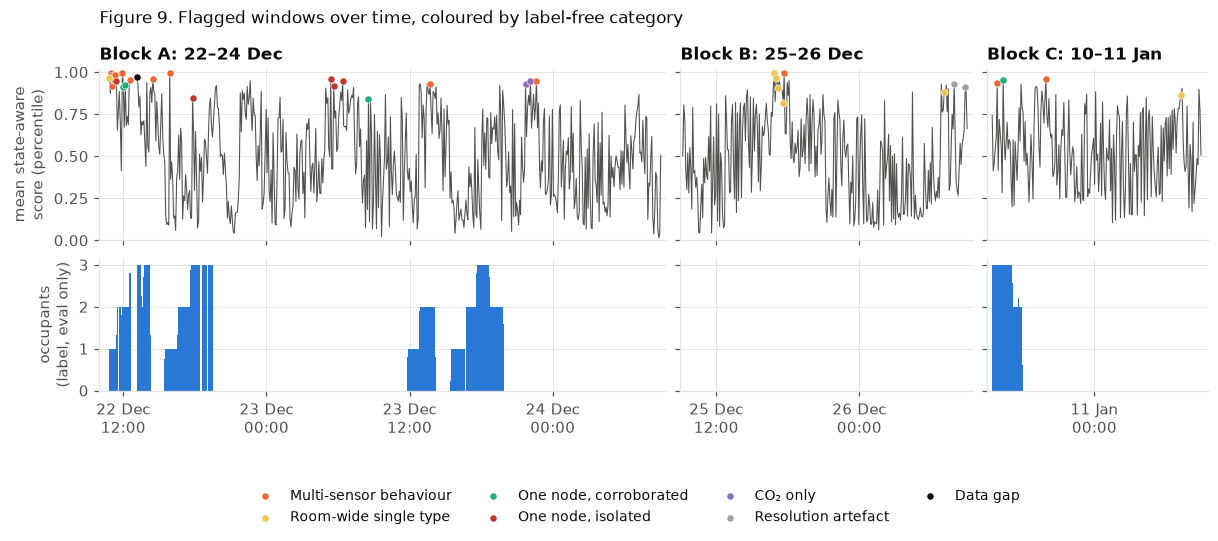

In [56]:
CAT_COL = {"Multi-sensor behaviour": C_ORANGE, "Room-wide single type": "#f2c14e",
           "One node, corroborated": C_AQUA, "One node, isolated": "#c0392b", "CO₂ only": "#8e6bbf",
           "Resolution artefact": C_GREY, "Data gap": INK}
fig, axes = plt.subplots(2, 3, figsize=(13, 3.8), sharey="row",
                         gridspec_kw={"width_ratios": widths, "height_ratios": [1.3, 1], "wspace": 0.04, "hspace": 0.12})
score = A_pct[STATE_SCORES].mean(axis=1)
for j, (a, b, title) in enumerate(blocks):
    a = pd.Timestamp(a)
    b = pd.Timestamp(b)

    m = (W["start"] >= a) & (W["start"] <= b)
    for _, g in W[m].groupby("segment"):
        axes[0, j].plot(g["start"], score[g.index], color=INK2, linewidth=0.7)
    for cat in CATS:
        mm = m & (W["anomaly_category"] == cat)
        axes[0, j].scatter(W.loc[mm, "start"], score[mm], s=22, color=CAT_COL[cat], zorder=3,
                           label=cat if j == 0 else None, edgecolor="white", linewidth=0.4)
    axes[1, j].bar(W.loc[m, "start"], W_lab.loc[m, "occ_mean"], width=pd.Timedelta(minutes=5),
                   color=C_BLUE, linewidth=0, align="edge")
    for ax in axes[:, j]:
        ax.set_xlim(a, b); ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
    axes[0, j].set_title(title); axes[0, j].tick_params(labelbottom=False)
axes[0, 0].set_ylabel("mean state-aware\nscore (percentile)"); axes[0, 0].set_ylim(0, 1.02)
axes[1, 0].set_ylabel("occupants\n(label, eval only)"); axes[1, 0].set_yticks([0, 1, 2, 3])
fig.legend(loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.24), fontsize=9)
fig.suptitle("Figure 9. Flagged windows over time, coloured by label-free category", x=0.125, ha="left", fontsize=11, y=1.02)
fig.savefig(f"{FIG_DIR}/fig9_anomaly_timeline.png"); plt.show()

### 4.7 Overall Findings and Limitations

The anomaly-detection analysis identified 35 potentially unusual windows using the state-aware consensus approach. Comparing global and state-aware detection demonstrated that the reference population influences which observations are considered unusual. Sensor-deviation analysis further showed that unusual observations involved different sensor features rather than one consistently dominant measurement.

Comparison with occupancy labels showed a higher anomaly rate during occupied windows (8.59%) than empty windows (2.13%). Transition windows also showed a higher anomaly rate (10.00%), although their small sample size limits the strength of this finding.

These results suggest that unusual sensor behaviour may be associated with room usage. However, the analysis cannot establish that flagged observations represent confirmed occupancy changes or faulty sensors. The limited recording periods, missing occupancy information in some recording segments and absence of direct sensor-health measurements restrict the conclusions. Therefore, detected anomalies should be treated as candidates for further investigation rather than confirmed faults.

# Section 5 – Arrival and Departure Detection

## 5.1 Overview and Analytical Objectives

This section investigates whether changes in room sensor readings can identify potential arrival and departure events without using occupancy labels during detection. The analysis uses the original 30-second-resolution sensor recordings to preserve temporal information that would be lost through five-minute aggregation.

The investigation follows these principles:

- **Temporal resolution:** Event detection uses the original 30-second sensor recordings. The group's existing five-minute clusters are attached only for descriptive linkage with RQ3; clustering is not repeated here.
- **Evaluation benchmark:** The primary benchmark consists of eight annotated whole-room occupancy transitions (empty to occupied or occupied to empty), rather than the 27 individual occupancy-count changes. Occupancy labels are used only after detection for evaluation and annotated visualisations.
- **Complete date coverage:** All seven recorded calendar dates are included in the evaluation, including dates with no annotated transitions. Unmatched detections on these dates count as false positives.
- **Detection approach:** The analysis uses causal and trailing sensor activity, direction-aware one-to-one event matching within ±1, ±2 and ±5-minute tolerances, and leave-date-out fitting of Sound and CO₂ thresholds.
- **Event timing:** Estimated event time is distinguished from confirmation time. In particular, departure confirmation requires at least 15 minutes of subsequent quiet activity.
- **Interpretation:** Results are treated cautiously because the benchmark contains only eight whole-room transitions. The analysis does not establish generalisable superiority of one detector over another.

The stored results include Fusion AND (7 true positives, 3 false positives and 1 false negative; F1 = 0.778) and filtered PIR (7 true positives, 5 false positives and 1 false negative; F1 = 0.700) at a ±2-minute matching tolerance. These results are checked against regression assertions in the notebook.

In [57]:
# Section 5 (re)defines the names below. If any already exist (e.g. inside the merged group notebook), they will be overwritten.
_S5_NAMES = ['df','raw','T','ALL','Z','X','M','P','Q','N','occ','e','g','cl','wl',
             'OUT','FIG','LAB','SND','ROOT','DATA_PATH','HOLD_MIN','GAP_SEC','delays','AUDIT']
_clash = [n for n in _S5_NAMES if n in globals()]
if _clash:
    print('WARNING: existing names will be overwritten by Section 5:', _clash)

## 5.2 Data and Dependencies

| Component | Description |
|---|---|
| Raw dataset | `Occupancy_Estimation.csv`, located beside the notebook or under `data/` |
| Cluster assignments | `data/results/clusters_k5.csv` |
| Cluster file columns | `segment`, `win`, `start`, `cluster`, `cluster_name`, `dist_to_centroid` |
| Required packages | NumPy, pandas, SciPy, Matplotlib and IPython |
| Previous-section dependencies | None required for standalone execution; `W` may optionally be used for a read-only consistency check |
| Results output | `data/results/section5_version6/` |
| Figure output | `figures/section5_version6/` |

**Execution:** Open the notebook from the packaged project directory, restart the kernel and run all cells in order.

In [58]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import beta
from IPython.display import display

pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110   # global setting (previously set in the figures cell)

ROOT = Path.cwd()
DATA_CANDIDATES = [ROOT/'Occupancy_Estimation.csv', ROOT/'data'/'Occupancy_Estimation.csv']
DATA_PATH = next((p for p in DATA_CANDIDATES if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place Occupancy_Estimation.csv beside this notebook or under data/')
OUT = Path('data/results/section5_version6'); FIG = Path('figures/section5_version6')
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

LAB = 'Room_Occupancy_Count'; SND = [f'S{i}_Sound' for i in range(1, 5)]
HOLD_MIN = 15; GAP_SEC = 300

raw = pd.read_csv(DATA_PATH)
required = ['Date', 'Time', LAB, 'S5_CO2', 'S6_PIR', 'S7_PIR'] + SND
missing = set(required) - set(raw)
assert not missing, f'Missing columns: {missing}'
df = raw.copy()
df['ts'] = pd.to_datetime(df['Date'].astype(str).str.replace('/', '-', regex=False) + ' ' + df['Time'].astype(str),
                          format='%Y-%m-%d %H:%M:%S')
df = df.sort_values('ts').reset_index(drop=True)
assert not df.ts.duplicated().any(), 'Duplicate timestamps need explicit resolution'
df['segment'] = (df.ts.diff().dt.total_seconds() > GAP_SEC).cumsum().astype(int)
df['date'] = df.ts.dt.date
ALL_DATES = sorted(df.date.unique())

print('Dataset:', DATA_PATH, '| shape:', df.shape, '| contiguous segments:', df.segment.nunique())
display(df.groupby('segment').ts.agg(['min', 'max', 'count']))

Dataset: /Users/kirtan/Professional/Queens University/Data mineing/Assignment - 1 /Notebook and prepared data/Final/data/Occupancy_Estimation.csv | shape: (10129, 22) | contiguous segments: 4


,min,max,count
segment,,,
0,2017-12-22 10:49:41,2017-12-22 12:42:31,216
1,2017-12-22 13:08:03,2017-12-24 09:10:50,5089
2,2017-12-25 09:11:42,2017-12-26 09:10:01,2779
3,2018-01-10 15:25:48,2018-01-11 09:00:09,2045


## 5.3 Data Preparation and Ground-Truth Events

The original 30-second sensor recordings are used to preserve the temporal characteristics of sensor responses. A new recording segment is created whenever the time gap between consecutive readings exceeds the specified `GAP_SEC` threshold.

For evaluation, all 27 annotated occupancy-count changes are extracted within the recording segments. However, the primary benchmark focuses on the eight whole-room transitions:

- **Arrival:** Empty to occupied.
- **Departure:** Occupied to empty.

This distinction prevents individual changes in occupant count from being treated as separate room-entry or room-exit events.

Occupancy annotations are retained exclusively for evaluation and visualisation. They are not used to determine detector activity or fit the detection thresholds.

In [59]:
e=df[['ts','segment','date',LAB]].copy()
e['count_before']=e.groupby('segment')[LAB].shift(); e['change']=e[LAB]-e.count_before
e=e[e.change.notna()&(e.change!=0)].rename(columns={LAB:'count_after'}).copy()
e['type']=np.where(e.change>0,'arrival','departure')
e['room_transition']=((e.count_before==0)&(e.count_after>0))|((e.count_before>0)&(e.count_after==0))
ALL=e.reset_index(drop=True); T=ALL[ALL.room_transition].reset_index(drop=True)
print(len(ALL),'count changes |',len(T),'room-level transitions:',T.type.value_counts().to_dict()); display(T[['ts','type','count_before','count_after']])
OCC_DATES=sorted(T.date.unique()); print('dates with room transitions:',OCC_DATES)

27 count changes | 8 room-level transitions: {'departure': 5, 'arrival': 3}


,ts,type,count_before,count_after
0,2017-12-22 14:15:58,departure,3.0,0
1,2017-12-22 15:25:24,arrival,0.0,1
2,2017-12-22 19:39:40,departure,3.0,0
3,2017-12-23 11:49:16,arrival,0.0,1
4,2017-12-23 14:10:11,departure,2.0,0
5,2017-12-23 15:26:46,arrival,0.0,1
6,2017-12-23 19:52:16,departure,2.0,0
7,2018-01-10 17:57:27,departure,2.0,0


dates with room transitions: [datetime.date(2017, 12, 22), datetime.date(2017, 12, 23), datetime.date(2018, 1, 10)]


## 5.4 Label-Free Event Detection

The event-detection approach combines sensor activity indicators and temporal persistence rules. Detection is performed without using occupancy labels.

In [60]:
def prepare(d,fit_mask,causal):
    x=d.copy(); x['snd']=x[SND].mean(axis=1); x['pir']=x[['S6_PIR','S7_PIR']].max(axis=1)
    s=x.snd[fit_mask]; lo=s[s<=s.quantile(.5)]; base=lo.median(); sig=1.4826*(lo-base).abs().median()
    thr=base+max(4*sig,0.02)
    def persist(b):
        n=b.astype(int).groupby(x.segment).transform(lambda v:v.rolling(7,center=not causal,min_periods=1).sum())
        return b&(n>=2)
    x['snd_act']=persist(x.snd>thr); x['pir_act']=persist(x.pir>0)
    x['fus_or']=x.snd_act|x.pir_act; x['fus_and']=x.snd_act&x.pir_act
    x['co2_d5']=x.groupby('segment')['S5_CO2'].diff(10)
    c=x.co2_d5[fit_mask].dropna(); cthr=max(10,3*1.4826*(c-c.median()).abs().median())
    return x,thr,cthr

def activity_events(x,col,hold,method):
    out=[]
    for seg,g in x.groupby('segment'):
        t0,t1=g.ts.iloc[0],g.ts.iloc[-1]; ts=g.ts[g[col]].reset_index(drop=True)
        for i,t in enumerate(ts):
            pre=(t-(ts[i-1] if i>0 else t0)).total_seconds()/60
            post=((ts[i+1] if i<len(ts)-1 else t1)-t).total_seconds()/60
            if pre>=hold:  out.append((seg,t,'arrival',pre,method,t))
            if post>=hold: out.append((seg,t,'departure',post,method,t+pd.Timedelta(minutes=hold)))
    return pd.DataFrame(out,columns=['segment','detected_time','event_type','detection_score','method','confirm_time'])

def co2_events(x,thr,refractory=10):
    out=[]
    for seg,g in x.groupby('segment'):
        v=g.co2_d5.values; ts=g.ts.values; last={'arrival':None,'departure':None}
        for i in range(1,len(v)):
            if np.isnan(v[i]) or np.isnan(v[i-1]): continue
            for typ,c in (('arrival',v[i]>=thr>v[i-1]),('departure',v[i]<=-thr<-v[i-1])):
                if c and (last[typ] is None or (ts[i]-last[typ])/np.timedelta64(1,'m')>=refractory):
                    t=pd.Timestamp(ts[i]); out.append((seg,t,typ,abs(v[i]),'CO2',t)); last[typ]=ts[i]
    return pd.DataFrame(out,columns=['segment','detected_time','event_type','detection_score','method','confirm_time'])

def run_all(d,fit_mask,causal,hold=HOLD_MIN):
    x,thr,cthr=prepare(d,fit_mask,causal)
    det={'PIR':activity_events(x,'pir_act',hold,'PIR'),'Sound':activity_events(x,'snd_act',hold,'Sound'),
         'CO2':co2_events(x,cthr),'Fusion OR':activity_events(x,'fus_or',hold,'Fusion OR'),
         'Fusion AND':activity_events(x,'fus_and',hold,'Fusion AND')}
    return det,x,thr,cthr

ALLROWS=pd.Series(True,index=df.index)
det_off,X_off,thr_off,cthr_off=run_all(df,ALLROWS,causal=False)
det_cau,X_cau,thr_cau,cthr_cau=run_all(df,ALLROWS,causal=True)
print('Sound thr',round(thr_off,3),'| CO2 thr',round(cthr_off,1),'| 10 readings ≈',round(df.groupby('segment').ts.diff(10).dt.total_seconds().median()/60,2),'min')

Sound thr 0.082 | CO2 thr 10 | 10 readings ≈ 5.1 min


## 5.5 Evaluation Protocol

### 5.5.1 Primary Evaluation: Leave-Date-Out Threshold Fitting

The principal evaluation uses the causal detector, leave-date-out threshold fitting and all seven recorded dates.

For each recorded calendar date, the Sound and CO₂ thresholds are fitted using data from all other recorded dates. Detections timestamped within the target date are then evaluated against the annotated events.

Importantly, dates without annotated transitions are retained. Any unmatched detections on these dates contribute to the false-positive count rather than being excluded from evaluation.

The detector operates over uninterrupted recording segments. Some segments extend across midnight and may therefore use sensor history from an adjacent date. Consequently, this procedure represents an offline leave-date-out threshold-fitting evaluation, not a complete isolation of temporal context.

In [61]:
def match(pred,truth,tol):
    """Maximum number of type-aware matches, then least total absolute timestamp error."""
    pred=pred.reset_index(drop=True); truth=truth.reset_index(drop=True)
    n,m=len(pred),len(truth)
    matched=[]
    if n and m:
        # Cost < 1 for allowed pairs; choosing an unmatched dummy costs 2;
        # invalid pairs cost 1e6. Thus maximise matches before minimising time error.
        invalid=1e6
        mat=np.full((n,n+m),invalid,dtype=float)
        mat[:,m:]=2.0
        for i,p in enumerate(pred.itertuples()):
            for j,t in enumerate(truth.itertuples()):
                dt=abs((p.detected_time-t.ts).total_seconds())/60
                if p.segment==t.segment and p.event_type==t.type and dt<=tol:
                    mat[i,j]=dt/(tol+1) # strictly <1
        ii,jj=linear_sum_assignment(mat)
        matched=[(i,j) for i,j in zip(ii,jj) if j<m and mat[i,j]<1]
    tp=len(matched); fp=n-tp; fn=m-tp
    P=tp/n if n else 0.;R=tp/m if m else 0.;F=2*P*R/(P+R) if P+R else 0.
    err=[(pred.loc[i,'detected_time']-truth.loc[j,'ts']).total_seconds()/60 for i,j in matched]
    lag=[(pred.loc[i,'confirm_time']-truth.loc[j,'ts']).total_seconds()/60 for i,j in matched]
    return dict(TP=tp,FP=fp,FN=fn,Precision=P,Recall=R,F1=F,
                MedianErr_min=float(np.median(err)) if err else np.nan,
                ConfirmLag_min=float(np.median(lag)) if lag else np.nan)

def loo_detections(causal, evaluated_days=None):
    """Fit thresholds without each scored date, pool every prediction for scored dates."""
    days=ALL_DATES if evaluated_days is None else list(evaluated_days)
    pooled={}
    for day in days:
        fitted,*_=run_all(df,df.date!=day,causal)
        for name,events in fitted.items():
            pooled.setdefault(name,[]).append(events[events.detected_time.dt.date==day].copy())
    return {k:pd.concat(v,ignore_index=True).sort_values('detected_time').reset_index(drop=True) for k,v in pooled.items()}

det_loo_off=loo_detections(False)
det_loo_cau=loo_detections(True)
det_loo_event_dates_only=loo_detections(True,OCC_DATES) # diagnostic only: reproduces Version 3 omission
scen={'1 Offline in-sample (all dates)':det_off,
      '2 Causal in-sample (all dates)':det_cau,
      '3a Leave-date-out offline (all 7)':det_loo_off,
      '3b Leave-date-out causal (all 7)':det_loo_cau,
      'OLD 3 event dates only (biased FP)':det_loo_event_dates_only}
rows=[]
for sname,det in scen.items():
    for method,preds in det.items():
        for tol in (1,2,5):
            rows.append(dict(scenario=sname,method=method,tol_min=tol,n_detected=len(preds),**match(preds,T,tol)))
M=pd.DataFrame(rows)
M.to_csv(OUT/'event_metrics_all_dates.csv',index=False)
for name,evs in [('in_sample_offline',det_off),('in_sample_causal',det_cau),
                 ('leave_date_out_offline_all7',det_loo_off),('leave_date_out_causal_all7',det_loo_cau)]:
    pd.concat(evs.values(),ignore_index=True).to_csv(OUT/f'detected_events_{name}.csv',index=False)
T.to_csv(OUT/'ground_truth_room_transitions_EVALUATION_ONLY.csv',index=False)
ALL.to_csv(OUT/'all27_count_changes_EVALUATION_ONLY.csv',index=False)
print('Recorded dates:',[str(x) for x in ALL_DATES], '| event dates:',[str(x) for x in OCC_DATES])
print('PRIMARY — leave-date-out causal, ±2 min')
display(M[(M.scenario=='3b Leave-date-out causal (all 7)')&(M.tol_min==2)][['method','n_detected','TP','FP','FN','Precision','Recall','F1','MedianErr_min','ConfirmLag_min']].round(3).sort_values('F1',ascending=False))
print('Tolerance sensitivity (±1, ±2, ±5 min)')
display(M[M.method.isin(['PIR','Fusion AND'])].pivot_table(index=['scenario','method'],columns='tol_min',values='F1').round(3))

Recorded dates: ['2017-12-22', '2017-12-23', '2017-12-24', '2017-12-25', '2017-12-26', '2018-01-10', '2018-01-11'] | event dates: ['2017-12-22', '2017-12-23', '2018-01-10']
PRIMARY — leave-date-out causal, ±2 min


,method,n_detected,TP,FP,FN,Precision,Recall,F1,MedianErr_min,ConfirmLag_min
58,Fusion AND,10,7,3,1,0.700,0.875,0.778,0.517,15.0
46,PIR,12,7,5,1,0.583,0.875,0.700,0.517,15.5
55,Fusion OR,42,5,37,3,0.119,0.625,0.200,0.000,15.0
49,Sound,44,5,39,3,0.114,0.625,0.192,0.000,15.0
52,CO2,141,1,140,7,0.007,0.125,0.013,0.500,0.5


Tolerance sensitivity (±1, ±2, ±5 min)


tol_min                                            1      2      5
scenario                           method                         
1 Offline in-sample (all dates)    Fusion AND  0.667  0.778  0.889
                                   PIR         0.600  0.700  0.800
2 Causal in-sample (all dates)     Fusion AND  0.556  0.778  0.889
                                   PIR         0.500  0.700  0.800
3a Leave-date-out offline (all 7)  Fusion AND  0.667  0.778  0.889
                                   PIR         0.600  0.700  0.800
3b Leave-date-out causal (all 7)   Fusion AND  0.556  0.778  0.889
                                   PIR         0.500  0.700  0.800
OLD 3 event dates only (biased FP) Fusion AND  0.556  0.778  0.889
                                   PIR         0.556  0.778  0.889

In [62]:
rows=[]
for typ in ('arrival','departure'):
    for m in ('PIR','Fusion AND'):
        p=det_loo_cau[m]; r=match(p[p.event_type==typ].reset_index(drop=True),T[T.type==typ].reset_index(drop=True),2)
        rows.append(dict(type=typ,method=m,**r))
display(pd.DataFrame(rows).round(2))
rows=[]
for h in (10,15,20,30,45):
    for causal in (False,True):
        det,*_=run_all(df,ALLROWS,causal,hold=h)
        for m in ('PIR','Fusion AND'): rows.append(dict(hold_min=h,window='causal' if causal else 'offline',method=m,F1=match(det[m],T,5)['F1']))
display(pd.DataFrame(rows).pivot_table(index='hold_min',columns=['window','method'],values='F1').round(2))

,type,method,TP,FP,FN,Precision,Recall,F1,MedianErr_min,ConfirmLag_min
0,arrival,PIR,3,2,0,0.60,1.0,0.75,0.00,0.00
1,arrival,Fusion AND,3,1,0,0.75,1.0,0.86,0.00,0.00
2,departure,PIR,4,3,1,0.57,0.8,0.67,0.52,15.52
3,departure,Fusion AND,4,2,1,0.67,0.8,0.73,0.52,15.52


window       causal          offline      
method   Fusion AND   PIR Fusion AND   PIR
hold_min                                  
10             0.73  0.73       0.62  0.57
15             0.89  0.80       0.89  0.80
20             0.89  0.80       0.89  0.80
30             0.89  0.80       0.89  0.80
45             0.86  0.75       0.86  0.75

## 5.6 Which sensor responds first? (ties explicit)
Per true room transition (offline flags). **Arrival:** time from the true event to the first active reading (negative = already active before the label; window −2…+15 min; CO₂: first rise ≥ threshold, −2…+30 min). **Departure:** time of the *last* active reading relative to the event (±10 min; CO₂: first fall, −2…+30 min). Two sensors are a **tie** if within 31 s (one sampling step). `NaN` = no response. This uses true times to align responses; it is not part of the detector.

**Important:** CO₂ often generates unrelated threshold crossings (141 alarms at ±2-min evaluation). Its rank as an early responder is *not* credible evidence of faster response, especially for departures. Distinguish last activity before departure from true physical sensor latency.


In [63]:
def first_true(g,col,t,lo,hi):
    w=g[(g.ts>=t+pd.Timedelta(minutes=lo))&(g.ts<=t+pd.Timedelta(minutes=hi))&g[col]]
    return (w.ts.iloc[0]-t).total_seconds()/60 if len(w) else np.nan
def last_true(g,col,t,lo,hi):
    w=g[(g.ts>=t+pd.Timedelta(minutes=lo))&(g.ts<=t+pd.Timedelta(minutes=hi))&g[col]]
    return (w.ts.iloc[-1]-t).total_seconds()/60 if len(w) else np.nan
X=X_off.copy(); X['co2_up']=X.co2_d5>=cthr_off; X['co2_dn']=X.co2_d5<=-cthr_off
rows=[]
for _,ev in T.iterrows():
    g=X[X.segment==ev.segment]; t=ev.ts
    if ev.type=='arrival': r=dict(PIR=first_true(g,'pir_act',t,-2,15),Sound=first_true(g,'snd_act',t,-2,15),CO2=first_true(g,'co2_up',t,-2,30))
    else: r=dict(PIR=last_true(g,'pir_act',t,-10,10),Sound=last_true(g,'snd_act',t,-10,10),CO2=first_true(g,'co2_dn',t,-2,30))
    rows.append(dict(event_time=t,type=ev.type,**r))
delays=pd.DataFrame(rows)
def winner(r):
    v=r[['PIR','Sound','CO2']].astype(float); 
    if r['type']=='arrival': v=v.where(v>=-2); k=v.dropna()
    else: k=v.dropna().abs()
    if k.empty: return 'none'
    best=k.min(); w=list(k[k<=best+0.52].index); return '+'.join(w)
delays['first_responder']=delays.apply(winner,axis=1)
delays.to_csv(OUT/'sensor_response_delays.csv',index=False); display(delays.round(2))
print(delays.groupby('type').first_responder.value_counts())
print(delays.groupby('type')[['PIR','Sound','CO2']].agg(['median','count']).round(2))

/var/folders/0h/47l1qjhn3ljfnsz7_cjvrv4m0000gn/T/ipykernel_22069/3977382286.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  delays.to_csv(OUT/'sensor_response_delays.csv',index=False); display(delays.round(2))


,event_time,type,PIR,Sound,CO2,first_responder
0,2017-12-22 14:15:58,departure,1.02,7.65,-1.53,PIR+CO2
1,2017-12-22 15:25:24,arrival,0.00,0.00,24.00,PIR+Sound
2,2017-12-22 19:39:40,departure,-3.07,0.00,0.00,Sound+CO2
3,2017-12-23 11:49:16,arrival,-0.52,-0.52,NaN,PIR+Sound
4,2017-12-23 14:10:11,departure,0.52,0.52,5.10,PIR+Sound
5,2017-12-23 15:26:46,arrival,-0.50,-0.50,14.82,PIR+Sound
6,2017-12-23 19:52:16,departure,0.52,0.52,4.60,PIR+Sound
7,2018-01-10 17:57:27,departure,0.50,0.00,4.08,PIR+Sound


type       first_responder
arrival    PIR+Sound          3
departure  PIR+Sound          3
           PIR+CO2            1
           Sound+CO2          1
Name: count, dtype: int64
             PIR        Sound          CO2      
          median count median count median count
type                                            
arrival    -0.50     3  -0.50     3  19.41     2
departure   0.52     5   0.52     5   4.08     5


## 5.7 Supplementary: all 27 count changes (incl. changes while people stay inside)
A within-room change (e.g. 2→3) may not alter sensors much. Test: does a short-term sensor change occur near the true change **more often than at random occupied times**? Change = trailing 4-reading mean − preceding 4-reading mean (≈2 min each, within segment, past data only). A sensor "responds" if |change| ≥ its unlabelled 97.5th percentile within [−0.5, +2] min of the time. Null = 2000 random times drawn from occupied readings (labels only used to choose the null sample). **Lift** = hit rate at true events ÷ null hit rate.

In [64]:
rng=np.random.default_rng(0)
Z=df.copy(); Z['sound']=np.log1p(Z[SND].clip(lower=0)).mean(axis=1); Z['pir']=Z[['S6_PIR','S7_PIR']].mean(axis=1); Z['co2']=Z.S5_CO2.astype(float)
def chg(s): return s.rolling(4,min_periods=4).mean()-s.shift(4).rolling(4,min_periods=4).mean()
cut={}
for k in ['sound','pir','co2']:
    Z[k+'_c']=Z.groupby('segment')[k].transform(chg); cut[k]=Z[k+'_c'].abs().quantile(.975)
    Z[k+'_hit']=Z[k+'_c'].abs()>=cut[k]
def hit(seg,t,k):
    w=Z[(Z.segment==seg)&(Z.ts>=t-pd.Timedelta(seconds=30))&(Z.ts<=t+pd.Timedelta(minutes=2))]; return bool(w[k+'_hit'].any())
occ=Z[Z[LAB]>0].sample(2000,replace=True,random_state=0)
rows=[]
for grp,sub in (('room transitions (8)',ALL[ALL.room_transition]),('within-room changes (19)',ALL[~ALL.room_transition]),('all changes (27)',ALL)):
    for k in ['pir','sound','co2']:
        h=np.mean([hit(r.segment,r.ts,k) for r in sub.itertuples()])
        n=np.mean([hit(r.segment,r.ts,k) for r in occ.itertuples()])
        rows.append(dict(group=grp,sensor=k,hit_rate=h,null_rate=n,lift=h/n if n else np.nan))
S27=pd.DataFrame(rows); S27.to_csv(OUT/'all27_response_vs_null.csv',index=False); display(S27.round(2))

,group,sensor,hit_rate,null_rate,lift
0,room transitions (8),pir,0.62,0.34,1.82
1,room transitions (8),sound,0.62,0.26,2.40
2,room transitions (8),co2,0.25,0.16,1.58
3,within-room changes (19),pir,0.63,0.34,1.84
4,within-room changes (19),sound,0.47,0.26,1.82
5,within-room changes (19),co2,0.26,0.16,1.66
6,all changes (27),pir,0.63,0.34,1.83
7,all changes (27),sound,0.52,0.26,1.99
8,all changes (27),co2,0.26,0.16,1.64


## 5.8 Figures

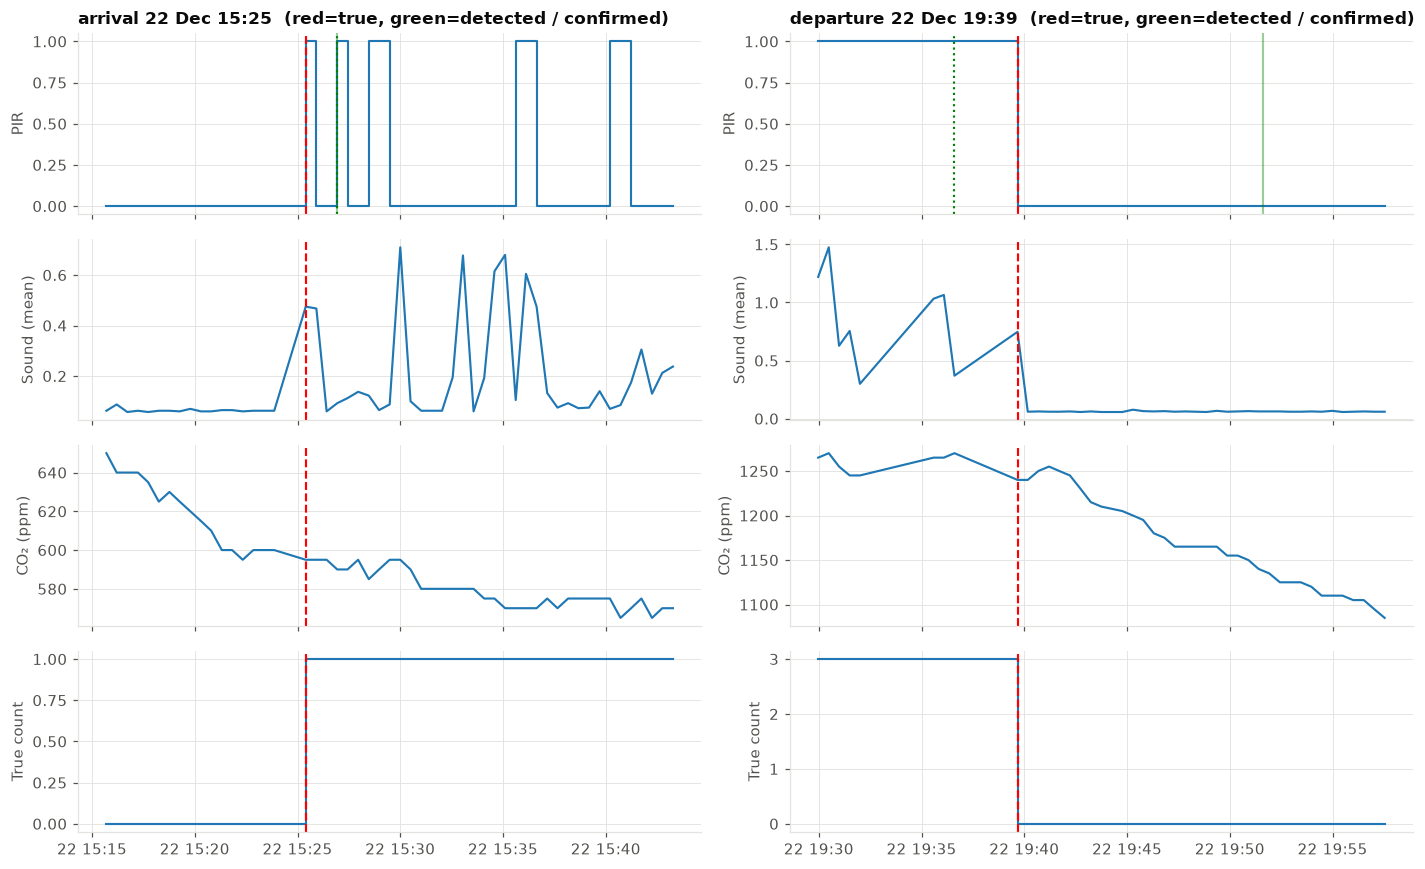

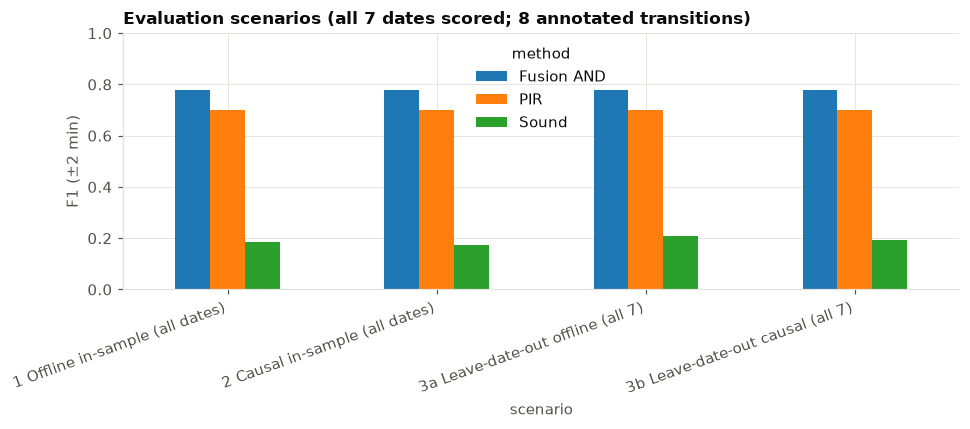

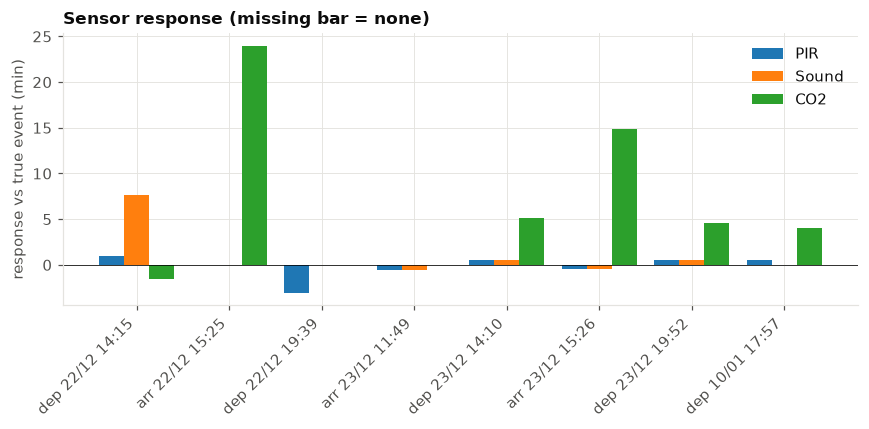

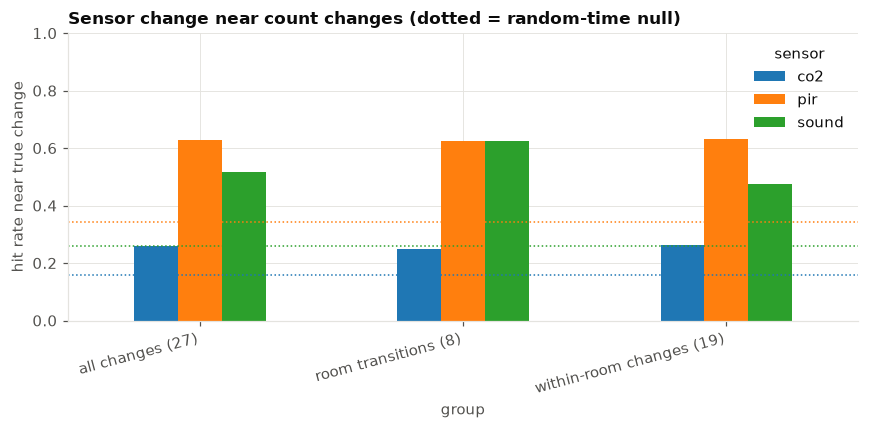

In [65]:
plt.rcParams['figure.dpi']=110
# Fig 1: example arrival + departure with sensors, causal Fusion AND detections
fig,axs=plt.subplots(4,2,figsize=(13,8),sharex='col')
for c,i in enumerate([1,2]):
    ev=T.iloc[i]; t=ev.ts; g=X_cau[(X_cau.ts>=t-pd.Timedelta(minutes=10))&(X_cau.ts<=t+pd.Timedelta(minutes=18))&(X_cau.segment==ev.segment)]
    for ax,(col,lab) in zip(axs[:,c],[('pir','PIR'),('snd','Sound (mean)'),('S5_CO2','CO₂ (ppm)'),(LAB,'True count')]):
        (ax.step(g.ts,g[col],where='post') if col in('pir',LAB) else ax.plot(g.ts,g[col])); ax.axvline(t,color='r',ls='--'); ax.set_ylabel(lab)
    pd_=det_cau['Fusion AND']; pd_=pd_[(pd_.detected_time>=g.ts.min())&(pd_.detected_time<=g.ts.max())&(pd_.segment==ev.segment)]
    for r in pd_.itertuples(): axs[0,c].axvline(r.detected_time,color='g',ls=':'); axs[0,c].axvline(r.confirm_time,color='g',ls='-',alpha=.4)
    axs[0,c].set_title(f'{ev.type} {t:%d %b %H:%M}  (red=true, green=detected / confirmed)')
fig.tight_layout(); fig.savefig(f'{FIG}/fig1_event_timeline.png',dpi=150); plt.show()
# Fig 2: performance by scenario
P=M[(M.tol_min==2)&(M.method.isin(['PIR','Fusion AND','Sound']))&(M.scenario!='OLD 3 event dates only (biased FP)')].pivot(index='scenario',columns='method',values='F1')
ax=P.plot.bar(figsize=(9,4)); ax.set_ylim(0,1); ax.set_ylabel('F1 (±2 min)'); ax.set_title('Evaluation scenarios (all 7 dates scored; 8 annotated transitions)'); plt.xticks(rotation=20,ha='right'); plt.tight_layout()
plt.savefig(f'{FIG}/fig2_performance_scenarios.png',dpi=150); plt.show()
# Fig 3: sensor responses
fig,ax=plt.subplots(figsize=(8,4)); xs=np.arange(len(delays)); w=.27
for k,(s,cl) in enumerate(zip(['PIR','Sound','CO2'],['tab:blue','tab:orange','tab:green'])): ax.bar(xs+(k-1)*w,delays[s],w,label=s,color=cl)
ax.set_xticks(xs); ax.set_xticklabels([f"{r.type[:3]} {r.event_time:%d/%m %H:%M}" for r in delays.itertuples()],rotation=45,ha='right')
ax.set_ylabel('response vs true event (min)'); ax.axhline(0,color='k',lw=.5); ax.legend(); ax.set_title('Sensor response (missing bar = none)'); plt.tight_layout()
plt.savefig(f'{FIG}/fig3_sensor_response.png',dpi=150); plt.show()
# Fig 4: all-27 lift
Q=S27.pivot(index='group',columns='sensor',values='hit_rate'); N=S27[S27.group=='all changes (27)'].set_index('sensor').null_rate
ax=Q.plot.bar(figsize=(8,4)); 
for i,(k,v) in enumerate(N.items()): ax.axhline(v,color=['C0','C1','C2'][['co2','pir','sound'].index(k)],ls=':',lw=1)
ax.set_ylim(0,1); ax.set_ylabel('hit rate near true change'); ax.set_title('Sensor change near count changes (dotted = random-time null)'); plt.xticks(rotation=15,ha='right'); plt.tight_layout()
plt.savefig(f'{FIG}/fig4_all27_vs_null.png',dpi=150); plt.show()

## Interpreting the corrected Version 6 findings

**Critical correction:** Prior Version 3 left out predictions from 4 calendar dates with no recorded room-transition events. In the **7-date complete scoring**, PIR changes from 7 TP / 3 FP / 1 FN (F1 0.778) to **7 TP / 5 FP / 1 FN (F1 0.700)**. Fusion AND remains **7 TP / 3 FP / 1 FN (F1 0.778)**. This is a *small apparent improvement* from two fewer false positives, **not evidence of universally superior fusion**.

**Main conclusion:** PIR+Sound AND detects some room-level transitions from unlabelled sensor activity. The 8 target events are not all 27 changes of person count. These detection counts represent offline event timestamp estimates, with confirmation at least 15 minutes after a departure. 1/2/5-minute tolerance is a reporting choice; sensitivity is provided. Extremely small sample, time dependence, uncertain reference annotations, and within-dataset model design preclude a generalised accuracy claim.

**Reference-label conflicts:** A false positive that coincides with noticeable sound and PIR activity while occupancy is labelled zero is a **sensor/annotation disagreement**. It still counts as FP under the reference labels; it does *not* establish that an unrecorded person entered. The near-missed departure on 22 Dec is separately investigated at ±5 min, not reclassified at ±2 min.

**Sensor response caveat:** PIR/Sound timestamp ties cannot identify a unique fastest device. CO₂ often changes later but no causal timing is proven. A change near a labelled event is not proof of its physical cause. The integration with Kirtan's K-means remains descriptive; ensure the cluster CSV provenance matches the final group pipeline.


## 5.9 Accuracy uncertainty, per-day failures and timestamps

Because this is a very small event benchmark, report **exact binomial 95% intervals** for observed precision (TP / predicted) and recall (TP / annotated events). These intervals are descriptive and assume trials are independent (an unrealistic simplification with time series), **not** guarantees of future performance. Inspect false positives and missed transitions; do not hide them. Separately record earliest `confirm_time` for prospective deployments.


In [66]:
def clopper_pearson(successes,total,alpha=.05):
    if total==0:return (np.nan,np.nan)
    return (0.0 if successes==0 else beta.ppf(alpha/2,successes,total-successes+1),
            1.0 if successes==total else beta.ppf(1-alpha/2,successes+1,total-successes))
primary=M[(M.scenario=='3b Leave-date-out causal (all 7)')&(M.tol_min==2)].copy()
primary['P_95_lo'],primary['P_95_hi']=zip(*[clopper_pearson(int(r.TP),int(r.TP+r.FP)) for r in primary.itertuples()])
primary['R_95_lo'],primary['R_95_hi']=zip(*[clopper_pearson(int(r.TP),int(r.TP+r.FN)) for r in primary.itertuples()])
primary.to_csv(OUT/'primary_metrics_with_uncertainty.csv',index=False)
display(primary[['method','TP','FP','FN','Precision','P_95_lo','P_95_hi','Recall','R_95_lo','R_95_hi','F1']].round(3))

def audit_event_matching(pred,truth,tol=2):
    # Assign globally under the same matching objective, expose matched and unmatched rows.
    p=pred.reset_index(drop=True);t=truth.reset_index(drop=True); n,m=len(p),len(t)
    mat=np.full((n,n+m),1e6,dtype=float);mat[:,m:]=2.
    for i,a in enumerate(p.itertuples()):
        for j,b in enumerate(t.itertuples()):
            diff=abs((a.detected_time-b.ts).total_seconds())/60
            if a.segment==b.segment and a.event_type==b.type and diff<=tol:mat[i,j]=diff/(tol+1)
    ii,jj=linear_sum_assignment(mat) if n and m else ([],[])
    pairs={int(i):int(j) for i,j in zip(ii,jj) if j<m and mat[i,j]<1}
    records=[]
    for i,r in p.iterrows():
        j=pairs.get(i)
        records.append({'status':'TP' if j is not None else 'FP','predicted_time':r.detected_time,'confirm_time':r.confirm_time,
                        'type':r.event_type,'true_time':t.loc[j,'ts'] if j is not None else pd.NaT,
                        'time_error_min':(r.detected_time-t.loc[j,'ts']).total_seconds()/60 if j is not None else np.nan,
                        'confirm_lag_min':(r.confirm_time-t.loc[j,'ts']).total_seconds()/60 if j is not None else np.nan})
    for j,r in t.iterrows():
        if j not in pairs.values():records.append({'status':'FN','predicted_time':pd.NaT,'confirm_time':pd.NaT,'type':r.type,'true_time':r.ts,'time_error_min':np.nan,'confirm_lag_min':np.nan})
    return pd.DataFrame(records)
AUDIT=audit_event_matching(det_loo_cau['Fusion AND'],T)
AUDIT.to_csv(OUT/'fusion_and_event_audit.csv',index=False)
print('Event-by-event audit (primary method):');display(AUDIT)
print('Performance by held-out event date (tiny denominators):')
perday=[]
for day in OCC_DATES:
    sub=T[T.ts.dt.date==day]
    for name in ['PIR','Fusion AND']:
        pred=det_loo_cau[name]; pred=pred[pred.detected_time.dt.date==day]
        perday.append({'date':str(day),'method':name,'n_true':len(sub),'n_pred':len(pred),**match(pred,sub,2)})
DAY=pd.DataFrame(perday);DAY.to_csv(OUT/'metrics_by_held_out_day.csv',index=False);display(DAY.round(3))


,method,TP,FP,FN,Precision,P_95_lo,P_95_hi,Recall,R_95_lo,R_95_hi,F1
46,PIR,7,5,1,0.583,0.277,0.848,0.875,0.473,0.997,0.700
49,Sound,5,39,3,0.114,0.038,0.246,0.625,0.245,0.915,0.192
52,CO2,1,140,7,0.007,0.000,0.039,0.125,0.003,0.527,0.013
55,Fusion OR,5,37,3,0.119,0.040,0.256,0.625,0.245,0.915,0.200
58,Fusion AND,7,3,1,0.700,0.348,0.933,0.875,0.473,0.997,0.778


Event-by-event audit (primary method):


,status,predicted_time,confirm_time,type,true_time,time_error_min,confirm_lag_min
0,TP,2017-12-22 14:16:59,2017-12-22 14:31:59,departure,2017-12-22 14:15:58,1.016667,16.016667
1,TP,2017-12-22 15:26:56,2017-12-22 15:26:56,arrival,2017-12-22 15:25:24,1.533333,1.533333
2,FP,2017-12-22 19:36:36,2017-12-22 19:51:36,departure,NaT,NaN,NaN
3,TP,2017-12-23 11:49:16,2017-12-23 11:49:16,arrival,2017-12-23 11:49:16,0.000000,0.000000
4,TP,2017-12-23 14:10:42,2017-12-23 14:25:42,departure,2017-12-23 14:10:11,0.516667,15.516667
5,FP,2017-12-23 14:43:53,2017-12-23 14:43:53,arrival,NaT,NaN,NaN
6,FP,2017-12-23 14:44:54,2017-12-23 14:59:54,departure,NaT,NaN,NaN
7,TP,2017-12-23 15:26:46,2017-12-23 15:26:46,arrival,2017-12-23 15:26:46,0.000000,0.000000
8,TP,2017-12-23 19:52:47,2017-12-23 20:07:47,departure,2017-12-23 19:52:16,0.516667,15.516667
9,TP,2018-01-10 17:57:27,2018-01-10 18:12:27,departure,2018-01-10 17:57:27,0.000000,15.000000


Performance by held-out event date (tiny denominators):


,date,method,n_true,n_pred,TP,FP,FN,Precision,Recall,F1,MedianErr_min,ConfirmLag_min
0,2017-12-22,PIR,3,3,2,1,1,0.667,0.667,0.667,1.275,8.775
1,2017-12-22,Fusion AND,3,3,2,1,1,0.667,0.667,0.667,1.275,8.775
2,2017-12-23,PIR,4,6,4,2,0,0.667,1.000,0.800,0.258,7.758
3,2017-12-23,Fusion AND,4,6,4,2,0,0.667,1.000,0.800,0.258,7.758
4,2018-01-10,PIR,1,1,1,0,0,1.000,1.000,1.000,0.500,15.500
5,2018-01-10,Fusion AND,1,1,1,0,0,1.000,1.000,1.000,0.000,15.000


## 5.10 Baseline and model comparison (replacing the weak shifted-time control)

A randomly shifted event-time null is almost guaranteed to give F1≈0 for sparse events at ±2 min. It is not a meaningful competing detector. We therefore compare a very simple **raw-PIR activity/quiet rule** (any PIR activation; no 2-of-7 persistence) with the production-style PIR and the PIR+Sound AND rule. Each method uses the same 15-minute quiet hold and is evaluated over **all 7 dates**. This baseline has no learnable sensor threshold and does not require fitting on occupancy labels. Results are exploratory because the model family and hold time were designed with knowledge of the data.


,method,n_detected,TP,FP,FN,Precision,Recall,F1
1,PIR,12,7,5,1,0.583,0.875,0.700
4,Fusion AND,10,7,3,1,0.700,0.875,0.778
7,Raw PIR (no persistence),19,6,13,2,0.316,0.750,0.444


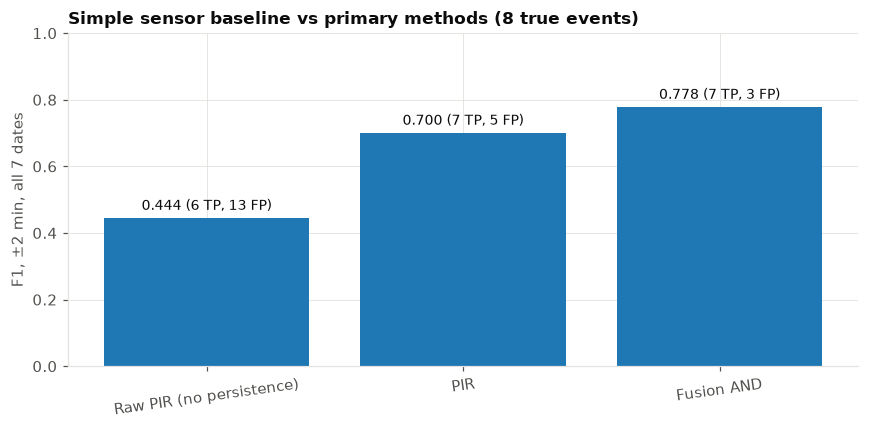

In [67]:
# Simple baseline: raw PIR on/off, no persistence; detects activity beginning or ending after a long quiet interval.
BASE_RAW= df.copy()
BASE_RAW['pir_raw']=(BASE_RAW[['S6_PIR','S7_PIR']].max(axis=1)>0)
raw_pir=activity_events(BASE_RAW,'pir_raw',HOLD_MIN,'Raw PIR (no persistence)')
BASELINE=pd.DataFrame([
    dict(method='Raw PIR (no persistence)',tol_min=tol,n_detected=len(raw_pir),**match(raw_pir,T,tol))
    for tol in (1,2,5)
])
BASELINE.to_csv(OUT/'simple_raw_pir_baseline.csv',index=False)
main_base = pd.concat([
    M[(M.scenario=='3b Leave-date-out causal (all 7)') & M.method.isin(['PIR','Fusion AND'])],
    BASELINE.assign(scenario='Baseline (raw PIR, all 7 dates)')
],ignore_index=True)
main_base.to_csv(OUT/'baseline_vs_primary.csv',index=False)
display(main_base[main_base.tol_min==2][['method','n_detected','TP','FP','FN','Precision','Recall','F1']].round(3))
fig,ax=plt.subplots(figsize=(8,4))
sel=main_base[main_base.tol_min==2].set_index('method').reindex(['Raw PIR (no persistence)','PIR','Fusion AND'])
ax.bar(range(len(sel)),sel.F1)
ax.set_xticks(range(len(sel)),sel.index,rotation=8)
ax.set_ylim(0,1);ax.set_ylabel('F1, ±2 min, all 7 dates')
ax.set_title('Simple sensor baseline vs primary methods (8 true events)')
for j,r in enumerate(sel.itertuples()):ax.text(j,r.F1+.025,f'{r.F1:.3f} ({r.TP} TP, {r.FP} FP)',ha='center',fontsize=9)
fig.tight_layout();fig.savefig(FIG/'fig5_raw_pir_baseline.png',dpi=180);plt.show()


## 5.10.1 Link to clusters (RQ3 integration)

If the shared notebook has already exported `data/results/clusters_k5.csv`, attach 5-minute room-state cluster names at the sensor event windows (no retraining here). This is **descriptive triangulation only**: the clusters themselves were estimated on the dataset, and this does not validate event detection. When the file is absent, report a clear skip rather than fabricate cluster relationships.


In [68]:
# Version 6: use the group-supplied clusters verbatim (never fit/re-label K-Means here).
# The notebook is still runnable standalone; within the merged group notebook, also compare to W.
cluster_candidates = [Path('data/results/clusters_k5.csv'), Path('clusters_k5.csv')]
cluster_file = next((p for p in cluster_candidates if p.exists()), None)
if cluster_file is None:
    raise FileNotFoundError('The group-provided clusters_k5.csv is required for Version 6. Put it under data/results/.')
cl = pd.read_csv(cluster_file, parse_dates=['start'])
needed = {'segment','win','start','cluster','cluster_name','dist_to_centroid'}
assert needed.issubset(cl.columns), f'Missing group cluster columns: {needed-set(cl.columns)}'
assert cl[['segment','win']].duplicated().sum() == 0, 'Duplicate group cluster window IDs'
assert len(cl) == 1044, f'Unexpected cluster window count: {len(cl)} (expected 1044 for this dataset)'
assert cl.cluster.nunique() == 5, 'Expected five group-derived clusters'
assert cl.start.notna().all(), 'Unparseable group cluster timestamps'
assert cl.groupby('segment').start.apply(lambda s:s.is_monotonic_increasing).all()
if 'W' in globals() and isinstance(W,pd.DataFrame) and {'segment','win','start','cluster','cluster_name'}.issubset(W.columns):
    group_check = W[['segment','win','start','cluster','cluster_name']].copy()
    file_check = cl[['segment','win','start','cluster','cluster_name']].copy()
    group_check['start']=pd.to_datetime(group_check['start'])
    group_check=group_check.sort_values(['segment','win']).reset_index(drop=True)
    file_check=file_check.sort_values(['segment','win']).reset_index(drop=True)
    pd.testing.assert_frame_equal(group_check,file_check,check_dtype=False)
    print('PASS: supplied cluster file exactly matches W from Section 7.4–7.8 of group notebook')
else:
    print('Standalone mode: cluster schema and window keys verified; full W comparison occurs in merged group notebook.')
print('Source of cluster assignments:',cluster_file,'| windows:',len(cl),'| clusters:',cl.cluster.value_counts().sort_index().to_dict())
# Link each detection to its actual 5-minute window by group segment AND window index.
# This avoids treating a nonexistent/low-fill window as a valid state.
segment_starts = df.groupby('segment').ts.min()
events6 = det_loo_cau['Fusion AND'].sort_values('detected_time').copy()
events6['win'] = [int((r.detected_time-segment_starts.loc[r.segment]).total_seconds()//300) for r in events6.itertuples()]
attached = events6.merge(cl[['segment','win','start','cluster','cluster_name','dist_to_centroid']],
                         on=['segment','win'],how='left',validate='many_to_one')
attached['window_age_min']=(attached.detected_time-attached.start).dt.total_seconds()/60
attached['has_group_cluster']=attached.cluster.notna()
assert (attached.window_age_min.dropna()>=0).all() and (attached.window_age_min.dropna()<5.001).all()
attached.to_csv(OUT/'v6_detected_events_with_official_group_clusters.csv',index=False)
print('Group cluster attached to',int(attached.has_group_cluster.sum()),'/',len(attached),'detected events.')
display(pd.crosstab(attached.event_type,attached.cluster_name,dropna=False))
# For descriptive context, sample the windows containing t-7.5 and t+7.5 min.
# Use actual group window IDs, without nearest-neighbour substitution across missing windows.
links=[]
cl_index=cl.set_index(['segment','win'])
for r in events6.itertuples():
    ss=segment_starts.loc[r.segment]
    def state_at(target):
        wn=int((target-ss).total_seconds()//300)
        idx=(int(r.segment),wn)
        return cl_index.loc[idx,'cluster_name'] if idx in cl_index.index else None
    links.append({'estimated_event_time':r.detected_time,'event_type':r.event_type,'segment':r.segment,
                  'cluster_7_5min_before':state_at(r.detected_time-pd.Timedelta(minutes=7.5)),
                  'cluster_7_5min_after':state_at(r.detected_time+pd.Timedelta(minutes=7.5))})
LINK6=pd.DataFrame(links)
LINK6['changed_cluster']=(LINK6.cluster_7_5min_before.notna() & LINK6.cluster_7_5min_after.notna() &
                           LINK6.cluster_7_5min_before.ne(LINK6.cluster_7_5min_after))
LINK6.to_csv(OUT/'v6_official_group_cluster_before_after.csv',index=False)
print('Descriptive room-state changes:');display(LINK6)
print('Important: clustering uses overlapping sensor data. This comparison is descriptive, NOT independent model validation.')


PASS: supplied cluster file exactly matches W from Section 7.4–7.8 of group notebook
Source of cluster assignments: data/results/clusters_k5.csv | windows: 1044 | clusters: {0: 82, 1: 545, 2: 88, 3: 216, 4: 113}
Group cluster attached to 9 / 10 detected events.


cluster_name,"Busy: high light, CO₂ rising",Occupied: moderate activity,NaN
event_type,,,
arrival,0,4,0
departure,3,2,1


Descriptive room-state changes:


,estimated_event_time,event_type,segment,cluster_7_5min_before,cluster_7_5min_after,changed_cluster
0,2017-12-22 14:16:59,departure,1,"Busy: high light, CO₂ rising","Recently vacated: dark, CO₂ falling",True
1,2017-12-22 15:26:56,arrival,1,"Recently vacated: dark, CO₂ falling",Occupied: moderate activity,True
2,2017-12-22 19:36:36,departure,1,"Busy: high light, CO₂ rising","Recently vacated: dark, CO₂ falling",True
3,2017-12-23 11:49:16,arrival,1,Empty: daylight only,Occupied: moderate activity,True
4,2017-12-23 14:10:42,departure,1,"Busy: high light, CO₂ rising","Recently vacated: dark, CO₂ falling",True
5,2017-12-23 14:43:53,arrival,1,"Recently vacated: dark, CO₂ falling",Occupied: moderate activity,True
6,2017-12-23 14:44:54,departure,1,"Recently vacated: dark, CO₂ falling",Occupied: moderate activity,True
7,2017-12-23 15:26:46,arrival,1,"Recently vacated: dark, CO₂ falling",Occupied: moderate activity,True
8,2017-12-23 19:52:47,departure,1,"Busy: high light, CO₂ rising","Recently vacated: dark, CO₂ falling",True
9,2018-01-10 17:57:27,departure,3,Occupied: moderate activity,"Recently vacated: dark, CO₂ falling",True


Important: clustering uses overlapping sensor data. This comparison is descriptive, NOT independent model validation.


## 5.10.2 poster handoff

**Preferred comparison:** all 7 recorded dates, causal leave-date-out sensor-threshold fitting. Note that only 3 dates contained any of the 8 fully empty/occupied reference transitions. Score every detector alert from all 7 dates. Report the **2-minute primary** and **5-minute sensitivity** side by side, plus a simple raw-PIR baseline.

**Poster text (verified again in the results table below):** Among 8 labelled whole-room transitions, Fusion AND identified 7 within ±2 min, with 3 unmatched alerts (P=0.70, R=0.875, F1=0.778). PIR alone found 7 with 5 unmatched alerts (P=0.583, R=0.875, F1=0.700), after correctly counting alerts on all 7 dates. At ±5 min, Fusion AND matched all 8 (F1=0.889). These are exploratory retrospective timestamp scores; departure confirmation requires ≥15 quiet minutes. Some unmatched alerts coincide with sensor activity despite a zero-occupancy label, not verified annotation faults. Do not generalise these small counts.

**RQ3 coordination:** Link events to existing 5-minute clusters and to Person 4 anomaly results, provided those are supplied by the team. The optional cluster join is not an independent validation. Confirm cluster-file seed, features, standardisation and label mapping against Kirtan's actual notebook before using the plot.


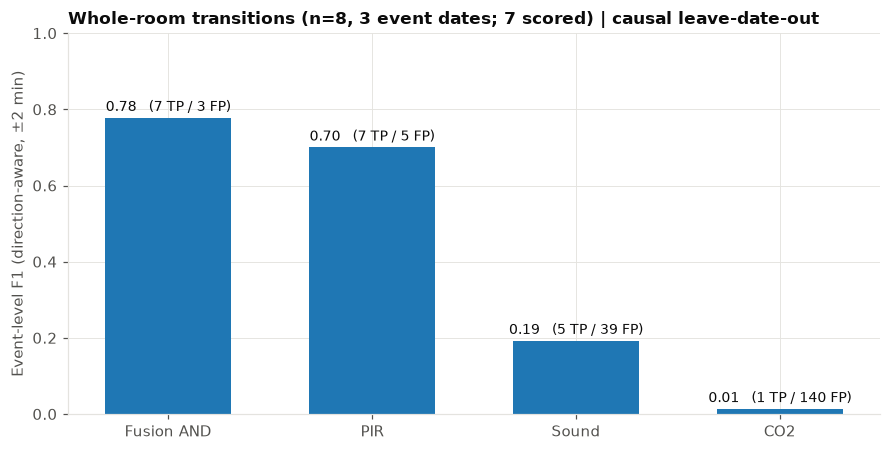

VERSION 6 COMPLETED — CSV: /Users/kirtan/Professional/Queens University/Data mineing/Assignment - 1 /Notebook and prepared data/Final/data/results/section5_version6  | Figures: /Users/kirtan/Professional/Queens University/Data mineing/Assignment - 1 /Notebook and prepared data/Final/figures/section5_version6


In [69]:
# One clean poster panel comparing *primary* methods, with event denominators visible.
sub=primary[primary.method.isin(['PIR','Sound','CO2','Fusion AND'])].set_index('method').loc[['Fusion AND','PIR','Sound','CO2']]
fig,ax=plt.subplots(figsize=(8.2,4.2))
xp=np.arange(len(sub)); bars=ax.bar(xp,sub.F1,width=.62)
for i,r in enumerate(sub.itertuples()):
    ax.text(i,r.F1+.018,f'{r.F1:.2f}   ({r.TP} TP / {r.FP} FP)',ha='center',fontsize=9)
ax.set_xticks(xp,sub.index,rotation=0);ax.set_ylim(0,max(1,sub.F1.max()+.12))
ax.set_ylabel('Event-level F1 (direction-aware, ±2 min)')
ax.set_title('Whole-room transitions (n=8, 3 event dates; 7 scored) | causal leave-date-out')
fig.tight_layout();fig.savefig(FIG/'fig6_primary_poster_performance.png',dpi=220);plt.show()
print('VERSION 6 COMPLETED — CSV:', OUT.resolve(),' | Figures:',FIG.resolve())


## 5.10.3 Forensic audit of unmatched alerts and near-misses

List *all* unmatched events. For any suspicious sensor activity under an occupancy label of zero, report the raw PIR and Sound readings and closest reference transition. **Keep the FP classification:** the available data cannot prove an annotation error. The December 22 ~19:36 versus ~19:39 departure is a tolerance-sensitive near miss, not a hit at ±2 min.


In [70]:
# Use independently audited 1:1 assignment; retain all-date false positives.
AUDIT5=audit_event_matching(det_loo_cau['Fusion AND'],T,5)
AUDIT5.to_csv(OUT/'fusion_and_audit_5min.csv',index=False)
AUDIT.to_csv(OUT/'fusion_and_audit_2min.csv',index=False)
print('2-minute event audit:');display(AUDIT.sort_values(['status','predicted_time'],na_position='last'))
print('5-minute event audit:');display(AUDIT5.groupby('status').size())
fp=AUDIT[AUDIT.status=='FP'].copy()
rows=[]
for r in fp.itertuples():
    nearest=df.iloc[(df.ts-r.predicted_time).abs().argsort()[:1]].iloc[0]
    reference=T[T.segment==nearest.segment]
    near=(reference.ts-r.predicted_time).abs().dt.total_seconds()/60
    rows.append({'predicted_time':r.predicted_time,'estimated_type':r.type,
                 'label_count_at_nearest_reading':int(nearest[LAB]),
                 'pir_s6':float(nearest['S6_PIR']),'pir_s7':float(nearest['S7_PIR']),
                 'mean_sound_at_reading':float(nearest[SND].mean()),
                 'closest_true_transition_min':float(near.min()) if len(near) else np.nan,
                 'note':'Unmatched under recorded occupancy labels; not proof of actual person or faulty annotation'})
FP_FORENSIC=pd.DataFrame(rows)
FP_FORENSIC.to_csv(OUT/'false_positive_sensor_audit.csv',index=False)
print('Unmatched signal evidence (do not relabel as true events):');display(FP_FORENSIC)


2-minute event audit:


,status,predicted_time,confirm_time,type,true_time,time_error_min,confirm_lag_min
10,FN,NaT,NaT,departure,2017-12-22 19:39:40,NaN,NaN
2,FP,2017-12-22 19:36:36,2017-12-22 19:51:36,departure,NaT,NaN,NaN
5,FP,2017-12-23 14:43:53,2017-12-23 14:43:53,arrival,NaT,NaN,NaN
6,FP,2017-12-23 14:44:54,2017-12-23 14:59:54,departure,NaT,NaN,NaN
0,TP,2017-12-22 14:16:59,2017-12-22 14:31:59,departure,2017-12-22 14:15:58,1.016667,16.016667
1,TP,2017-12-22 15:26:56,2017-12-22 15:26:56,arrival,2017-12-22 15:25:24,1.533333,1.533333
3,TP,2017-12-23 11:49:16,2017-12-23 11:49:16,arrival,2017-12-23 11:49:16,0.000000,0.000000
4,TP,2017-12-23 14:10:42,2017-12-23 14:25:42,departure,2017-12-23 14:10:11,0.516667,15.516667
7,TP,2017-12-23 15:26:46,2017-12-23 15:26:46,arrival,2017-12-23 15:26:46,0.000000,0.000000
8,TP,2017-12-23 19:52:47,2017-12-23 20:07:47,departure,2017-12-23 19:52:16,0.516667,15.516667


5-minute event audit:


status
FP    2
TP    8
dtype: int64

Unmatched signal evidence (do not relabel as true events):


,predicted_time,estimated_type,label_count_at_nearest_reading,pir_s6,pir_s7,mean_sound_at_reading,closest_true_transition_min,note
0,2017-12-22 19:36:36,departure,3,1.0,1.0,0.3700,3.066667,Unmatched under recorded occupancy labels; not...
1,2017-12-23 14:43:53,arrival,0,1.0,0.0,0.3200,33.700000,Unmatched under recorded occupancy labels; not...
2,2017-12-23 14:44:54,departure,0,1.0,0.0,0.6325,34.716667,Unmatched under recorded occupancy labels; not...


## 5.10.4 Seven-date accountability and headline tolerance table

Every recorded date must be shown, including dates with zero true transitions. For days where the 15-minute hold uses readings across midnight, the event is attributed to the calendar date of its *estimated* timestamp. This makes the evaluation reproducible, but does not represent a live prospective date-by-date deployment.


**Unit of evaluation:** the 8 annotated whole-room transitions; each predicted arrival and departure counts separately. A brief unannotated burst may generate both an unmatched arrival and departure. An optional episode view can group that burst for interpretation but must **not** replace the primary event-level F1.


In [71]:
all_day_rows=[]
for day in ALL_DATES:
    truth=T[T.ts.dt.date==day]
    for method in ['PIR','Fusion AND','Sound','CO2']:
        pred=det_loo_cau[method];pred=pred[pred.detected_time.dt.date==day]
        all_day_rows.append(dict(date=str(day),method=method,n_truth=len(truth),n_detected=len(pred),**match(pred,truth,2)))
DAYS7=pd.DataFrame(all_day_rows)
DAYS7.to_csv(OUT/'seven_date_detection_accountability.csv',index=False)
display(DAYS7[DAYS7.method.isin(['PIR','Fusion AND'])][['date','method','n_truth','n_detected','TP','FP','FN']])
TOL=M[(M.scenario=='3b Leave-date-out causal (all 7)')&(M.method.isin(['Fusion AND','PIR']))]
display(TOL[['method','tol_min','TP','FP','FN','Precision','Recall','F1','ConfirmLag_min']].sort_values(['method','tol_min']).round(3))
TOL.to_csv(OUT/'poster_2min_5min_tolerance.csv',index=False)
assert (DAYS7[DAYS7.method=='PIR'].FP.sum()==match(det_loo_cau['PIR'],T,2)['FP'])
assert (DAYS7[DAYS7.method=='Fusion AND'].FP.sum()==match(det_loo_cau['Fusion AND'],T,2)['FP'])
assert match(det_loo_cau['PIR'],T,2)['FP']==5
assert match(det_loo_cau['Fusion AND'],T,2)['FP']==3
print('All-date evaluation checks PASS')


,date,method,n_truth,n_detected,TP,FP,FN
0,2017-12-22,PIR,3,3,2,1,1
1,2017-12-22,Fusion AND,3,3,2,1,1
4,2017-12-23,PIR,4,6,4,2,0
5,2017-12-23,Fusion AND,4,6,4,2,0
8,2017-12-24,PIR,0,0,0,0,0
9,2017-12-24,Fusion AND,0,0,0,0,0
12,2017-12-25,PIR,0,2,0,2,0
13,2017-12-25,Fusion AND,0,0,0,0,0
16,2017-12-26,PIR,0,0,0,0,0
17,2017-12-26,Fusion AND,0,0,0,0,0


,method,tol_min,TP,FP,FN,Precision,Recall,F1,ConfirmLag_min
57,Fusion AND,1,5,5,3,0.500,0.625,0.556,15.000
58,Fusion AND,2,7,3,1,0.700,0.875,0.778,15.000
59,Fusion AND,5,8,2,0,0.800,1.000,0.889,13.467
45,PIR,1,5,7,3,0.417,0.625,0.500,15.500
46,PIR,2,7,5,1,0.583,0.875,0.700,15.500
47,PIR,5,8,4,0,0.667,1.000,0.800,13.717


All-date evaluation checks PASS


### conclusions and integrity checklist

- All 7 dates scored (including zero-event dates): **yes**.
- Sensor thresholds held out by evaluated date: **yes**; fixed detector design is exploratory, not cross-validated.
- Labels used only in scoring/diagnostic figures, not in detection threshold fitting: **yes**.
- Event-estimate and confirmation timestamps kept separate: **yes**.
- ±2 min and ±5 min displayed together; unmatched active readings retained as FP: **yes**.
- All 27 changes versus 8 room transitions explicitly distinguished: **yes**.
- Full reproducibility: CSV, notebook, event audit and figure exports. **Check group file provenance and official assessment brief separately before submission.**


## 5.11 independent methodological audit (what changed and what did not)

**Primary result stays fixed:** all **7** recorded dates, causal sensor windows, threshold fitting without the scored calendar date, direction-aware one-to-one ±2-minute matching, **8** annotated whole-room transitions. Unmatched predictions on zero-transition dates count as false positives.

**Three distinct quantities must not be confused:** (a) an *estimated event timestamp* inferred from a sensor transition; (b) the later *confirmation timestamp*, which for a departure requires 15 minutes of quiet; (c) the **annotation interval** between the last old occupancy label and first new label when observations are missing.

The remaining analyses are **diagnostic/sensitivity analyses** only. They do not tune the detector on the reference annotations, do not alter the 7/3/1 primary counts, and do not claim to confirm an unrecorded entry.

In [72]:
# --- Integrity: re-check primary numbers against unfiltered 7-date predictions ---
assert len(ALL_DATES)==7 and len(ALL)==27 and len(T)==8
v6_main=[]
for method in ['Raw PIR (no persistence)','PIR','Fusion AND','Sound','CO2']:
    p=raw_pir if method.startswith('Raw ') else det_loo_cau[method]
    for tol in (1,2,5):
        v6_main.append({'method':method,'tolerance_min':tol,'n_predictions':len(p),**match(p,T,tol)})
V6_PRIMARY=pd.DataFrame(v6_main)
assert match(det_loo_cau['Fusion AND'],T,2)['TP']==7
assert match(det_loo_cau['Fusion AND'],T,2)['FP']==3
assert match(det_loo_cau['PIR'],T,2)['FP']==5
V6_PRIMARY.to_csv(OUT/'v6_primary_all7_tolerance_1_2_5.csv',index=False)
display(V6_PRIMARY[V6_PRIMARY.tolerance_min==2].round(3))
print('All 7 dates evaluated; primary confusion counts preserved.')

,method,tolerance_min,n_predictions,TP,FP,FN,Precision,Recall,F1,MedianErr_min,ConfirmLag_min
1,Raw PIR (no persistence),2,19,6,13,2,0.316,0.750,0.444,0.250,7.75
4,PIR,2,12,7,5,1,0.583,0.875,0.700,0.517,15.50
7,Fusion AND,2,10,7,3,1,0.700,0.875,0.778,0.517,15.00
10,Sound,2,44,5,39,3,0.114,0.625,0.192,0.000,15.00
13,CO2,2,141,1,140,7,0.007,0.125,0.013,0.500,0.50


All 7 dates evaluated; primary confusion counts preserved.


## 5.11.1 Two alarms versus one short activity episode (supplementary only)

A 2017-12-23 **14:43:53** arrival alarm followed by a **14:44:54** departure alarm overlaps a short activity burst while the occupancy count is labelled zero. The event-level benchmark legitimately counts **both unmatched predicted transitions** (one false arrival and one false departure). For *investigation workload*, these can be regarded as one contiguous **unmatched activity episode**. The number of false-alert episodes is descriptive and **must not be substituted into event-level Precision/F1**.

A possible interpretation is an unannotated presence, activity transmitted from outside the monitored space, sensor noise or a label issue; **the data alone cannot establish which**.

In [73]:
# Cluster only UNMATCHED Fusion AND alerts in the same segment within 2 minutes.
fp6=AUDIT[AUDIT.status=='FP'].copy().sort_values('predicted_time').reset_index(drop=True)
seg_lookup=df.set_index('ts')['segment']
fp6['segment']=fp6.predicted_time.map(seg_lookup)
fp6['delta_prev_min']=fp6.predicted_time.diff().dt.total_seconds()/60
join_previous=(fp6.segment.eq(fp6.segment.shift()) & fp6.delta_prev_min.le(2))
fp6['episode_id']=(~join_previous).cumsum()
episodes=fp6.groupby('episode_id',as_index=False).agg(
    start=('predicted_time','min'),end=('predicted_time','max'),
    number_of_unmatched_transition_alarms=('status','size'),
    event_types=('type',lambda z:', '.join(z))
)
episodes['duration_between_alarms_sec']=(episodes.end-episodes.start).dt.total_seconds()
fp6.to_csv(OUT/'v6_unmatched_alarm_episode_assignments.csv',index=False)
episodes.to_csv(OUT/'v6_false_alarm_episodes_descriptive.csv',index=False)
print('Primary unmatched transition alarms:',len(fp6),'| Descriptive unmatched alert episodes:',len(episodes))
display(episodes)
assert len(fp6)==3 and len(episodes)==2

Primary unmatched transition alarms: 3 | Descriptive unmatched alert episodes: 2


,episode_id,start,end,number_of_unmatched_transition_alarms,event_types,duration_between_alarms_sec
0,1,2017-12-22 19:36:36,2017-12-22 19:36:36,1,departure,0.0
1,2,2017-12-23 14:43:53,2017-12-23 14:44:54,2,"arrival, departure",61.0


## 5.11.2 Gap-aware annotation audit: do NOT silently turn a miss into a hit

For an occupancy-count change observed just after an acquisition gap, its physical transition could have occurred **anywhere between** the last observation with the old label and the first observation with the new label. We report that interval and whether a detector estimate lies at/near the interval boundary; this flags **time-label uncertainty**, not validated correctness. The main ±2-minute matching continues to use recorded annotation timestamps.

For the 2017-12-22 evening departure, the final recorded activity occurs at **19:36:36** and the new zero-occupancy annotation is at **19:39:40** (184 seconds apart). The estimated departure at 19:36:36 is at the **old-label boundary**; it is not logically proved to be inside an open interval following that old-label observation. Under a more lenient ±5-minute tolerance it does match. Both distinctions are documented.

In [74]:
g= df[['ts','segment',LAB]].copy()
g['previous_ts']=g.groupby('segment').ts.shift()
g['previous_count']=g.groupby('segment')[LAB].shift()
uncertain=g[(g[LAB]!=g.previous_count)&g.previous_count.notna()].copy()
uncertain['gap_sec']=(uncertain.ts-uncertain.previous_ts).dt.total_seconds()
uncertain['transition_type']=np.where(uncertain[LAB]>uncertain.previous_count,'arrival','departure')
trans_uncertain=uncertain[(((uncertain.previous_count==0)&(uncertain[LAB]>0))|((uncertain.previous_count>0)&(uncertain[LAB]==0)))].copy()
# Connect each reference event to its nearest same-direction predicted event within 5 minutes, for investigation only.
extra=[]
for _,r in trans_uncertain.iterrows():
    sub=det_loo_cau['Fusion AND']
    sub=sub[(sub.segment==r.segment)&(sub.event_type==r.transition_type)].copy()
    sub['signed_offset_min']=(sub.detected_time-r.ts).dt.total_seconds()/60
    sub=sub[sub.signed_offset_min.abs()<=5].sort_values('signed_offset_min',key=lambda z:z.abs())
    candidate=sub.iloc[0] if len(sub) else None
    extra.append({'annotation_ts':r.ts,'event_type':r.transition_type,'last_old_label_ts':r.previous_ts,
                  'annotation_gap_sec':r.gap_sec,'nearest_prediction_within_5min':candidate.detected_time if candidate is not None else pd.NaT,
                  'prediction_within_open_gap':bool(r.previous_ts<candidate.detected_time<=r.ts) if candidate is not None else False,
                  'prediction_at_old_label_boundary':bool(candidate.detected_time==r.previous_ts) if candidate is not None else False})
GAP_AUDIT=pd.DataFrame(extra)
GAP_AUDIT.to_csv(OUT/'v6_ground_truth_timestamp_uncertainty.csv',index=False)
display(GAP_AUDIT[GAP_AUDIT.annotation_gap_sec>90])

,annotation_ts,event_type,last_old_label_ts,annotation_gap_sec,nearest_prediction_within_5min,prediction_within_open_gap,prediction_at_old_label_boundary
1,2017-12-22 15:25:24,arrival,2017-12-22 15:23:52,92.0,2017-12-22 15:26:56,False,False
2,2017-12-22 19:39:40,departure,2017-12-22 19:36:36,184.0,2017-12-22 19:36:36,False,True


## 5.11.3 HOLD_MIN sensitivity on the **same primary benchmark**

The earlier hold sensitivity table only reported ±5-minute **in-sample** results. Here we repeat it with **causal sensor windows, leave-date-out Sound/CO₂ threshold fitting, all seven dates scored, and ±2 minutes**. This is still a *post-hoc sensitivity analysis* on the dataset used throughout development; it is **not** hyperparameter optimization or a fresh held-out test. The chosen `HOLD_MIN = 15` remains fixed for the headline result.

In [75]:
HOLD_VALUES=(10,15,20,30,45)
# Cache per-fold sensor activity; only post-processing needs repeating for each hold.
fold_x={}
for day in ALL_DATES:
    fold_x[day]=prepare(df,df.date!=day,True)[0]
sens=[]
for hold in HOLD_VALUES:
    for method,flag in [('PIR','pir_act'),('Fusion AND','fus_and')]:
        preds=[]
        for day,x in fold_x.items():
            p=activity_events(x,flag,hold,method)
            preds.append(p[p.detected_time.dt.date==day])
        p=pd.concat(preds,ignore_index=True)
        for tol in (2,5):
            sens.append({'hold_min':hold,'method':method,'tolerance_min':tol,'n_pred':len(p),**match(p,T,tol)})
HOLD_SENS=pd.DataFrame(sens)
HOLD_SENS.to_csv(OUT/'v6_hold_sensitivity_causal_leave_date_out_all7.csv',index=False)
display(HOLD_SENS[HOLD_SENS.tolerance_min==2][['hold_min','method','n_pred','TP','FP','FN','F1']].round(3))
assert (HOLD_SENS.query('hold_min==15 and method=="Fusion AND" and tolerance_min==2').iloc[0].F1 == match(det_loo_cau['Fusion AND'],T,2)['F1'])

,hold_min,method,n_pred,TP,FP,FN,F1
0,10,PIR,14,7,7,1,0.636
2,10,Fusion AND,14,7,7,1,0.636
4,15,PIR,12,7,5,1,0.700
6,15,Fusion AND,10,7,3,1,0.778
8,20,PIR,12,7,5,1,0.700
10,20,Fusion AND,10,7,3,1,0.778
12,30,PIR,12,7,5,1,0.700
14,30,Fusion AND,10,7,3,1,0.778
16,45,PIR,8,5,3,3,0.625
18,45,Fusion AND,6,5,1,3,0.714


## 5.11.4 Sensor response: direction and specificity matter

PIR and Sound response timings should be described as *sensor activity relative to labels*, not proven physical reaction times. The departure analysis uses **last active timestamps**, not first changes. The high CO₂ alarm rate (141 total) prevents a reliable claim that CO₂ was an equally fast departure sensor. For a clean poster-facing comparison, exclude CO₂ from any *fastest detector* ranking, while **retaining its standalone baseline performance and its measured values**. Avoid concluding that an unmatched zero-label activity confirms a label fault.

In [76]:
# A compact non-misleading sensor-response summary.
RESP_V6=delays[['event_time','type','PIR','Sound','CO2']].copy()
RESP_V6['PIR_vs_Sound']=np.select(
    [RESP_V6.PIR.isna()&RESP_V6.Sound.isna(),RESP_V6.PIR.isna(),RESP_V6.Sound.isna(),
     (RESP_V6.PIR-RESP_V6.Sound).abs()<=0.52,RESP_V6.PIR<RESP_V6.Sound],
    ['no detected response','Sound only','PIR only','indistinguishable at ~30s cadence','PIR earlier'],
    default='Sound earlier')
RESP_V6['CO2_caveat']='CO2 threshold crossings not used to declare fastest response'
RESP_V6.to_csv(OUT/'v6_response_interpretation_PIR_sound_CO2_caveat.csv',index=False)
display(RESP_V6)
print('PIR vs Sound (descriptive, not a prospective latency benchmark):',RESP_V6.groupby(['type','PIR_vs_Sound']).size().to_dict())

,event_time,type,PIR,Sound,CO2,PIR_vs_Sound,CO2_caveat
0,2017-12-22 14:15:58,departure,1.016667,7.650000,-1.533333,PIR earlier,CO2 threshold crossings not used to declare fa...
1,2017-12-22 15:25:24,arrival,0.000000,0.000000,24.000000,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
2,2017-12-22 19:39:40,departure,-3.066667,0.000000,0.000000,PIR earlier,CO2 threshold crossings not used to declare fa...
3,2017-12-23 11:49:16,arrival,-0.516667,-0.516667,NaN,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
4,2017-12-23 14:10:11,departure,0.516667,0.516667,5.100000,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
5,2017-12-23 15:26:46,arrival,-0.500000,-0.500000,14.816667,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
6,2017-12-23 19:52:16,departure,0.516667,0.516667,4.600000,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
7,2018-01-10 17:57:27,departure,0.500000,0.000000,4.083333,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...


PIR vs Sound (descriptive, not a prospective latency benchmark): {('arrival', 'indistinguishable at ~30s cadence'): 3, ('departure', 'PIR earlier'): 2, ('departure', 'indistinguishable at ~30s cadence'): 3}


## 5.11.5 Results for the poster — pre-specified primary versus exploratory diagnostics

**Main statement:** On all 7 dates and **8 annotated whole-room transitions** (3 arrivals, 5 departures), causal ±2-min detection returned **Fusion AND: 7 TP, 3 FP, 1 FN (F1 = 0.778)** and **PIR alone: 7 TP, 5 FP, 1 FN (F1 = 0.700)**. The difference of two false predictions is too small to establish generalizable superiority. At ±5 min, the additional 2017-12-22 departure is matched, but this does not remove uncertainty from its 184-s annotation gap.

**What not to claim:** detection of all 27 occupancy-count changes, independent external validation, real-time 0-minute exit detection, verified missing person labels, or CO₂ as an equally prompt response channel. The leave-date-out exercise estimates only sound/CO₂ thresholds on other dates; the pipeline structure was iteratively developed with knowledge of this dataset. Departure confirmation requires **15 min quiet**.

**Episode secondary analysis:** 3 unmatched transition alarms correspond to 2 temporally separated unmatched alert episodes (one of which comprises arrival/departure alarms around 14:44). This does **not** change primary FP/F1.

**RQ3 link:** compare detected room transitions with team-established 5-minute K-Means clusters, strictly as descriptive convergence rather than independent verification.

**Confidence intervals:** precision and recall intervals are wide because only eight transitions were annotated. The expected value is in the critical interpretation, not just in a CSV.

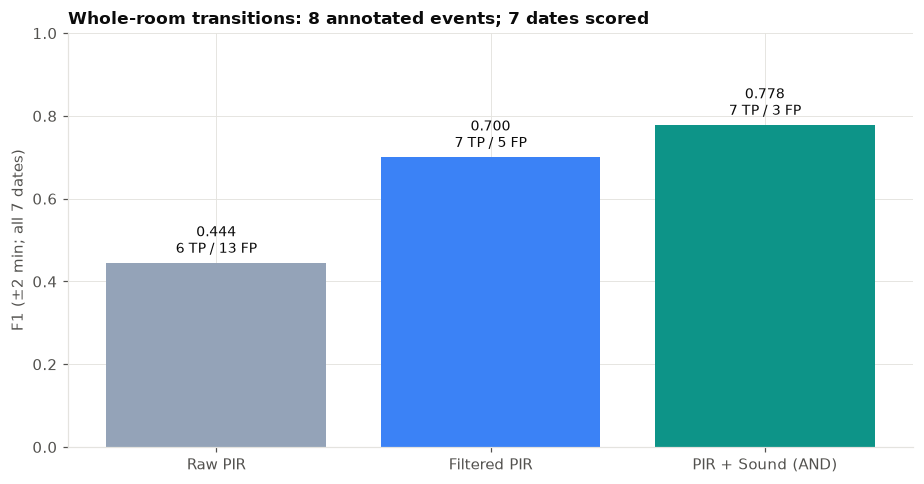

Final consistency: {'main_2min': {'TP': 7, 'FP': 3, 'FN': 1, 'Precision': 0.7, 'Recall': 0.875, 'F1': 0.7777777777777777, 'MedianErr_min': 0.5166666666666667, 'ConfirmLag_min': 15.0}, 'main_5min': {'TP': 8, 'FP': 2, 'FN': 0, 'Precision': 0.8, 'Recall': 1.0, 'F1': 0.888888888888889, 'MedianErr_min': 0.25833333333333336, 'ConfirmLag_min': 13.466666666666667}}


In [77]:
# Export a one-page summary table that can be pasted into the group poster.
poster=V6_PRIMARY[V6_PRIMARY.method.isin(['PIR','Fusion AND','Raw PIR (no persistence)']) & V6_PRIMARY.tolerance_min.isin([2,5])].copy()
poster=poster[['method','tolerance_min','n_predictions','TP','FP','FN','Precision','Recall','F1','ConfirmLag_min']]
poster.to_csv(OUT/'v6_poster_headline_table.csv',index=False)
fig,ax=plt.subplots(figsize=(8.5,4.5))
a=V6_PRIMARY[V6_PRIMARY.tolerance_min==2].set_index('method').loc[['Raw PIR (no persistence)','PIR','Fusion AND']]
bars=ax.bar(range(3),a.F1,color=['#94a3b8','#3b82f6','#0d9488'])
ax.set_xticks(range(3),['Raw PIR','Filtered PIR','PIR + Sound (AND)'])
ax.set_ylim(0,1); ax.set_ylabel('F1 (±2 min; all 7 dates)')
ax.set_title('Whole-room transitions: 8 annotated events; 7 dates scored')
for bar,row in zip(bars,a.itertuples()):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.025,f'{row.F1:.3f}\n{row.TP} TP / {row.FP} FP',ha='center',fontsize=9)
fig.tight_layout();fig.savefig(FIG/'fig7_v6_primary_methods_all_dates.png',dpi=200);plt.show()
print('Final consistency:',{'main_2min':match(det_loo_cau['Fusion AND'],T,2),'main_5min':match(det_loo_cau['Fusion AND'],T,5)})

## 5.12 Final group-integration handoff — Arash Ansarimehr

The joined K-Means states are **directly sourced from the supplied final Group 5 notebook**, not independently re-created. Section 5 is an **RQ2 supporting analysis** for the wider RQ3 interpretation of room states/anomalies. Anomaly observations supplied by Person 4 should be joined separately; none are invented here.

**Claims safe for poster:** 7/8 whole-room transitions detected within ±2 minutes; 3 false event alarms on 7 days; AND F1=.778 vs filtered PIR F1=.700; ±5-minute F1=.889; departure confirmations need ≥15 minutes; only 8 room-level events among 27 occupancy-count changes. Sensor responses are descriptive, and CO₂ is not an effective sharp event-clock under these rules. Confidence bounds are broad.

**Not safe to claim:** we detect every individual entering/leaving, measured sensor-caused lags, external generalisation, a verified annotation error, or proof the cluster link independently validates the detector.

Group poster ready metrics:


,method,tolerance_min,n_reference_room_events,dates_scored,TP,FP,FN,Precision,Recall,F1,ConfirmLag_min
0,Raw PIR (no persistence),2,8,7,6,13,2,0.316,0.750,0.444,7.750
1,Raw PIR (no persistence),5,8,7,7,12,1,0.368,0.875,0.519,11.933
2,PIR,2,8,7,7,5,1,0.583,0.875,0.700,15.500
3,PIR,5,8,7,8,4,0,0.667,1.000,0.800,13.717
4,Sound,2,8,7,5,39,3,0.114,0.625,0.192,15.000
5,Sound,5,8,7,5,39,3,0.114,0.625,0.192,15.000
6,CO2,2,8,7,1,140,7,0.007,0.125,0.013,0.500
7,CO2,5,8,7,3,138,5,0.021,0.375,0.040,4.083
8,Fusion AND,2,8,7,7,3,1,0.700,0.875,0.778,15.000
9,Fusion AND,5,8,7,8,2,0,0.800,1.000,0.889,13.467


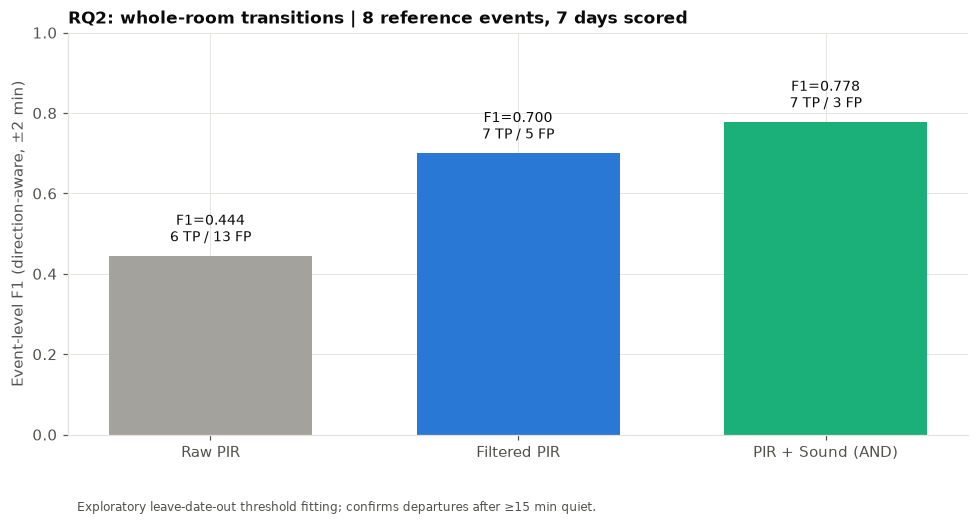

In [78]:
# Compact, fresh handoff exports: numbers below are recomputed from detections, not copied from markdown.
summary6=[]
for method in ['Raw PIR (no persistence)','PIR','Sound','CO2','Fusion AND']:
    predictions=raw_pir if method=='Raw PIR (no persistence)' else det_loo_cau[method]
    for tol in [2,5]:
        score=match(predictions,T,tol)
        summary6.append({'method':method,'tolerance_min':tol,
                         'n_reference_room_events':len(T),'dates_scored':len(ALL_DATES),
                         'n_predicted':len(predictions),**score})
HANDOFF6=pd.DataFrame(summary6)
HANDOFF6.to_csv(OUT/'v6_GROUP_POSTER_METRICS.csv',index=False)
print('Group poster ready metrics:')
display(HANDOFF6[['method','tolerance_min','n_reference_room_events','dates_scored','TP','FP','FN','Precision','Recall','F1','ConfirmLag_min']].round(3))
assert HANDOFF6.query('method=="Fusion AND" and tolerance_min==2').iloc[0][['TP','FP','FN']].tolist()==[7,3,1]
assert HANDOFF6.query('method=="PIR" and tolerance_min==2').iloc[0][['TP','FP','FN']].tolist()==[7,5,1]
assert HANDOFF6.query('method=="Fusion AND" and tolerance_min==5').iloc[0][['TP','FP','FN']].tolist()==[8,2,0]
fig, ax=plt.subplots(figsize=(9.0,4.9))
main=HANDOFF6.query('tolerance_min==2 and method in ["Raw PIR (no persistence)","PIR","Fusion AND"]').copy()
main=main.set_index('method').loc[['Raw PIR (no persistence)','PIR','Fusion AND']].reset_index()
colors=['#a3a29c','#2a78d6','#1baf7a']
bars=ax.bar(['Raw PIR','Filtered PIR','PIR + Sound (AND)'], main.F1, color=colors, width=.66)
for b,(_,r) in zip(bars,main.iterrows()):
    ax.text(b.get_x()+b.get_width()/2,b.get_height()+.025,
            f"F1={r.F1:.3f}\n{int(r.TP)} TP / {int(r.FP)} FP",ha='center',va='bottom',fontsize=9)
ax.set_ylim(0,1);ax.set_ylabel('Event-level F1 (direction-aware, ±2 min)')
ax.set_title('RQ2: whole-room transitions | 8 reference events, 7 days scored')
ax.text(0.01,-.19,'Exploratory leave-date-out threshold fitting; confirms departures after ≥15 min quiet.',
        transform=ax.transAxes,fontsize=8,color='#52514e')
fig.tight_layout();fig.savefig(FIG/'v6_GROUP_POSTER_primary_methods.png',dpi=250,bbox_inches='tight');plt.show()

## 6. Synthesis and Overall Findings

This section brings together the findings from data preparation, clustering, anomaly detection and arrival/departure analysis to address the overall research question: **Can unlabelled sensor readings reveal distinct room-usage patterns and unusual periods, and how can unusual room behaviour be distinguished from potential sensor faults?**

In [79]:
# Self-contained notebook data (no external CSVs or ZIPs needed).
# The archive below is the frozen source evidence from the group draft.
# It expands only into a temporary directory for this notebook run.
from pathlib import Path as _DataPath
import base64 as _b64, io as _io, zipfile as _zip, tempfile as _temp, shutil as _shutil

_EMBEDDED_ARCHIVE_B85 = (
    'P)h>@6aWAK2mlF;cU}KyzlZz10RS#H4gehh003lRbYU+~V`Fu2VQyo2Uqy3tX>DP2X>V>WV{>-2y-'
    'Sa7y^bC>&u^(+Ub;&)bvy_Vz=7NI1H&;K18KJh_8|X0ix+9>POW!Wqx;lXd!O_1SrjRXqNqpz`+xeM|K;mH{<nYrFJJ$p{_!9G%Rm2*uYc0~Ps9JT{7?0d|MS27*Z=2#!vBDOG5Hspe^'
    'LMVr+@ih|NZ}l{|*0Q@-H_3;{Ne(|Gnma{Ntbg-+%cZH@5%B|Mh?Thp&GM_>ceaFaPq-|M>U+`9J@!|M8#x`+xrb{_$_`f9-$%Z~9W<-zfcWwEj}pk4-;TeQEohEc^@(emei9-'
    'M5KfN~<qpznuB9*VpxZ#rua!@SCR}Cc)napR~E~r~118;!AZX?)p)Bj$$pLn1YfF$aVvYw_Z6D;ip}p*c-)F5H-'
    'T1hXn+svPK2LDM=6YqfCq77Z4yl|K~~!U}DTl=oP>%YYSirK*ef+DjhTr5&WD(=pU6KqS`{379uc&@&&`KAgo(yaXk>~+ki6}oo!OIxEhyIGYs>ioTvtme%2t7X932a`!}T|Ma+-'
    '&6A*V}=r7~G?myCpr^aXRkz<U7AK4!j=5jCk_5gCtceLpEFg{>!lZxEhlVF4<5EdZdgJwfSpN}y58w>z0|7}1S7(PPLl^NzJ?&o&IDGH2{$snkK&OW8=GbwHqQ~T4@*6xl|6-tDk-V7-'
    'G@i%}Ye=Qz$qu6?4Oi}!gO1&<O;#+0ZxAz50H_AAh2kee53mA7TlzCtxjhO=-R47=*ue^Dt$Q&m8-'
    '2ciU3>pMslxqepC}|poJ7#TQbPc0zo+T<zL`NvkM4Zo;_@nj4G`jXP{TM$qFkbY4c!w_01F|xvAe2SKoq0g|(MEFT8^ujxa6vJlctDtsS-'
    'N8Y$b=PZgJKJc?G_UV0A{;jsh{im(N=UbwhTF!8<n|=m(8_79Oo9=_+il03<rMM2mBjG{b+v%qbOq1^pE5V_QF+upGF{x^J~*s1WA=H1j4#7h<VbXIf(wzVE{=JFH;m|vJw~$7^GcgrX'
    'Vg#Ac-f8%Gsj|dAJ;|Y}-(FgP0$^0vV>|<IjY0gDcD)tCV7e;?gmSFHw_IBSI14<&9#0^brb-Oo}<2(Xe?QF(Em+QQSRY5GBdFs1j$i$sPuO73&eZ<|sy;pt#~)v09hO#X^)KjKAm0sV'
    '-F>#x6~EiTluxC`O;6n2-%mS-4}AbZv9*8ztOsHb(*9=XH$d%Qa;9Y?oB6FAEg2LNWcC-'
    '0ikt>XR;FsEoHWZ%~@ZkJixj0>da`+>bxTJt(w)Tv|UAU0g=NdE~eG#f_3~XFm3^IG||Q%UoKRF6qa3Q58;OE08>38X~n4G`Sc4YXAvup2X@<%+A>*g9sD<1~Fl-NoD#}O?+L_WeAlxT'
    'w2luj6c^TgZO8aEJK!RlW4P#E%*PMc&Z4+{3q{M6OdVGQTjH$I8ic)uA)6HUuUCrZ@I6{Xkkv_uP;&}ESxLs1B<%%+yaRI^7pueTNte^x}<%#CI&TGiMAN!X;Zuw?Q#7BBb1N=e#@e#<'
    '8QI}bS7Fo@itFx14E;$jqo)Gu?rBKcLc)Y-&G6B_-iGAI4VEQG)cWD>DVrX#mH_Y+nUWNwR1YO(KgTN%L`uWsrIxt1&<OcKn}#yn?Y1vlbC{F^=YdKfVkp7suU$i6Ie2Y<xd5wKW%N1Q'
    'BtXT<n01D?EUw3NmI>HumE+0Qi@&b@!T832}y~HRE%mcqMBRYw?<K{NVGyua)a1#YLxVZj+~M5-)}3xH%j7i)M6Gks*ovMRo=8ze-6@IPh5`DbpdiVS~``gd4nMB-Sow!sEJ8Z8))yb@'
    '9O1|4IjO*4b>M{qIx|Z2u-nE)!qf^E*d=;VRxtjV>M7s*hL*w?N#J#!rtHpaB8K2$-%_s@+s|fA}`+dXv3y8m!5E|GeSJ8sxR4&D%M6j)TO#>4&kN{!^E(ak?VOOtxno-'
    '#c76Mn{i6je5jO2PRI#w2r4(t#>qBe$~4|oln~w3a;d392(Di_jB7IVVr+3wb3;&-X$^7b8nF~h%d+7aAxaTSyC1zn2w(o*f!$;F9iM$aM=N$G(GrfUOAAZf5bg`@tYg11XH#6lZdrS-'
    'EzPtrj}}ndFNWqH)}bk?k(xsUF8Y`%EsU{7Q6+rP;Ru++k#hkEgst(+0wq(S$K*NCTj37d5cxbF3BnIoEUvTYt3I-rfJCnI(Eh@95gcU1fZmky*1|Sh3q-'
    'kMZHN2c?okrgc}5ga<sJ;Jd_lpqIXopFn^8JlCMYyi4N5Tu%ot-'
    'CMSX{W9}c?kYJ>)lsY!K46mxN%XQ9jO(k6jlk+{6Nav&kc4Q=Ih3PNQb0x|IcxqqsAW32COh!0=rN5PZ~k-Umhptfc)0fD;c01_Jz{dH$jFcK6%Oew$JZbk#<+pYc-hRQtSfYmSwU~V6'
    'V5p%v26g|VZw!%Mw(Ol;lt&g4z+L^C#5lm1yNu>SR?G!kBe4pt~V2qWuVawp=(wm}9MoAKi;X;oov88e4$27$t<~g=h*))A#GJ!FE?g0fxF^v8WDK`vg@;64Q{cNg?<yy}H3LH!2NJcR'
    'xvO8P15>7Rq#iR$}7kihcw7~~ffukfu|H_A_D2|If*!8eN$<Br8u6AWFmF;1a3}Y&o*^Inn3&9wQ`38NMt1%4IFN*_==St54##b;LU7{+@BKO4ibm-D8jT0D?=7Tn9!?Og-'
    'O8ID<U~IoH9AFYx8wkctqP|BIlcN}h7n(1(69-30@if>ct~Ri2KNU`{3zgNp5-UCrw-FbCHhCXm?8WtlwF;p`NE|3rs`^k>LX<A`ouXLRE0b)mOrm&?p+3ZVClawPBdm{Balv6kL90LZ'
    'D2MsR)tixo4L5PWcHJn}3%Z1_JIZ4uv1Q0|-'
    'r_Dm3C)S#1V#TSZW8INUsTB;cOo3h%Ee_A0!gW!CQ}e9Ijlk4SI}iLQfZ9W`+y+&{!_bCA3zLO941zYk5v@e9=#a>43{to#k%$cbb?}|V0*_X`gYh{+t-'
    '}9Iw;$Iho&!KGGLag4sHi>kt*oHIAs)XAP6Mcc0WA<p`wFZ`j;(UjA^7P6-Nyq?vBt(wY#hV#Bt$)#*0$?PL&4*CNEWk3~%NLMeFv&c!EOJ2e$-q?8W-~QYAKW%1R(ch{D!${b2-'
    '&jTgI|Mw<Af#SYr-?op_nSj{k;K2zkLiMdLU*I=hX4=2sWz$FN`vxtF?Iu7`{oPsE54h2Pm+3$yL5NGxtY|CKL7T8p~Y-'
    'a%^`Z}4IfJClCY)1<<VI^GYd;pUmNa}ioCLmOakcW%SPD=1Op0i++bO~W4aWR7G1p*31N1xN8dqxsUJ6=;1?g;d}X&}%Ws6bePpm^e{+7Lm6dGK`?mmxaI<>O8Hc&f|Q2hh%e9eh`tn?'
    'Sf{5%Fm<LJx=vWm<5|A`lz*bKEJebx3+B$`^I%3{Z?<rt|ui>yjY19(k*)b`a+<1`0FIX|8kZAwu32#^-'
    '!fGlUZS#~Chi5JYfmh^LcS@u@aJT&8W7oj@1~0*}oV9{`8qq5&avUEi2PST1k$5IKtLqJ@3RO*!H5u(ZZ$rRf$-'
    'C5_$!aWFDf$jbM7mK)|3IOn*GvHIdiu&b;0kP4vOzO7e}0LJXTT;r%mN}3hzU}-1A2u|&DX6Lzf(Wy{EPe$PFaVTY_JD+tP>}t9W=m~_ef?XNn-sUN)NNetba{;t4LSE(q7cFK1R8<g|'
    '#oQ2O0^F09Alg#G6v9+7I@x}p(xZjNj3V#%O@>f*zZY|ns}%s@sjN^SJQa}`0`e{LQBMab_g^D~P^i2iOn4xo>a?($r!ls0-'
    '8%@Mo9rM`AjGBii@!@hR}b+`dS#0<iqGYiR8^83ZuL?S44$}L0U)6_MSKDUTA}1)cW!}uywr3$_Tn}4(q8G&A(j4J&k8&%nl;&<G_MV;!8V{Ggeef=`{}FaVPbo$VhoBOn)_T?kF?u+X'
    '=tNW*8`&6#G@>El-7MO9YE-'
    '&mtX;5)dOLhp#lh7oOb9r_7_bHL5X`STp_p`AT$6~*NCeT`WCtgg4Gp*mmun9V3!~W>aMkIfH2%*LlD8OhbeU3TK>W)yWMIbfHe=m<Fah+M~#HuS@IZ_t&M7=-'
    'QE=H+*~dq6koj7!_R^Oqf#BqJx8*6u-'
    'aCL35vCQi~9<}*V!;St=jG#H1y>vH+5Q4!&igF8NI5mNR5+k0b;%2Ri4aYbkhof0|gM#3g+;+N`w$5&W+CIz*@&+c*h`qdm?}!R3(DlPvA4b5ri#bhZ9qW)fTrHq`=joBjGVN_X%K4Lg'
    '7{kDg>?$F-qK{lqguT5Goi+fhux!s79dz@x&TexwE97SVbqYQ_;2(ZS7WpvCG%1S@YR|lDH_eAEx+)<#9cRbF%SNuv5b4yRVQ)aCHF7Crh4Mq22a$K||NAu3(-'
    'SSFL!qz|i4XK8C%+nx|Ii{h<<~P%Vg2wjlP|H3q5#GKvfPc#aJtIhk#B!TcaJFnB;l<rK<nJvRdGs(=VW)u6d50W*X<>+^VKnR54lrmWUex8yc)*3fsWt!NYgxhPCra6rySS@(SM*tlx'
    '8Stp`6_n^>KA((qrIA_1beN4=u&@zDSdL{<|!<C>Opq(4FZ@Ey8FdU<Z9&CP|N>kwEIjd2oA5L;i&GF(Z77OlwpCG*6=eEl71ulSy{V*wxPq+<JT$5E4smR`;DaTIbQ#}YAH*#WILtM{'
    'Vk+SP*)`K9TkgqAn)gXrGZQ+|hi>HX8bn_IKO7qWmd|!)XU%vl*Qv}n=q%KiJq2N1Z7FKQLxgtbUJI2Wfu^-`r=Y6&3h7r<Thwns-'
    'z!f2eP!l`n(4n|(PUp~J5Wx!*E^tAJ5Q3`_ct4!j0J<n)^Ee@d6geUnga{&)yPBM(@lG=EwAP$EW1P~6p}zM$HHcyKI2)cc(3H3lN)XJ4M&w6P2@r{^M8kw=P!dI1JQJo?4V6(q5ihM5'
    'iAzQOoM<xh9Lp*1s0(O>;<m?Z8X97+9m*5T(dIg@;hI~=3B_I_3RR32Bj)nDMAPuO%IFD?P_(dP(u#{l8x&o_Ee2UzU1|47&!B|NQ!BomwHUD0hbzho?k)A!bttods5MuP5GCI~8EjID'
    'n`JJ-!o+=a`=sYaFk!04g8=iIj&O6qg0}&r#3ih-'
    '+Hg&02EpzNw#}>ebCeLX62c~2TQ2Jmf>C2^CneZ*pZhZ&%{}Rloj{loA~i}VnjLs1RhpU<BSd5O+e+=Yro#wvIngy1XUoxrr$O`FaxKHy3dU`n3In1x)eS~Q={uGO6wkGt9%X>=w(2lt'
    'ubTD~Pav$`D`GhPoLwr+im3h8Ne8a)5Q??6COpYgjZt4PV@;GaSb<ACu-F#Mr!ippt7#(lPbh&FSIL7Tmv~4MJ=laa(d8;l-'
    'Kb6&O_SjQ!`jto`DT{5s<)8Upx)2z(FvTnafzpyCNsOM+$^igshDLHr@auf64!VJlwuE+*tc9^4+(i|!xtI_5OZ;rXFXa7g1xf3<kj5X!XT>KK$#JQsyyUe&UfP#af_}mSTHaUQckLA`'
    'GtOPNBdpdp7ISiitkd@IN)TA1Lw#0-'
    '+>9r`G7WgD`I2TXC>UmN4Ph0;rHH{HfVUP1!vrrLcVt!*_x|6^@l@zuVmkrxdUK6lEF=~CX+{(g`2MPYl34d9BU^yfpDOe2`5R^8RzzCPlbonotX_dhKoHMO;o{QYlAYHlqs!pjyC25;'
    'Y3>-F8lD1b(%1U3Jg+Q7pv1YkC+o(*K*khwmFfD(u8wI4jM6+aWw6za55$;X0SGX+bW4LRQF-'
    '$N)y94x=!Fq22u9sP{krOFCmjRj{BKvCw_3?SQm$lad3ri$^hhlaob^tFjV`YQHyF0bI(0I#SDB4!*DhMe~md;*ZwdV$8-6IV1iq~xG(H}z(ycE-'
    'K3g0w763Jr`_;QU|a<g;{wK#Hb{08k)}#<F)QHCq}!4XFyW{4Jv@UJ=P(?z!c(nr4C5q^4qOHrVZfsi25zo62$Gt3iEe+xKxV!zqj)I-'
    'M6Lu8O0shl@Bk`V(y_L|mSs5eB$yxtw8#aa21X4qnj$_OIX_wD9r5u%wclnBFo}yob8T>XRxtUthoKX64PDN&qu~jRD=?`wf5AZW8;Fz!IwlpwHna;Jsk;4u*^BE#qb9SNX>%7j9bDW#'
    'fro4=?Sr$uxb^7_CGrgkMOzkF1o*^IfKgm0nv7R5y<(e$QaX*a><2u*HC?VZU}!EB%~dJOKEf!9%(zR%rQqI&kt$M*v6^prZ6<$sw8452?owke4^GZldl-YXF}apm>Jpg4+`lSpLA?J;'
    '<NXEh8H06+>~hPD3i{o2+{I-?p&ARLm=?vhD3J>-nhqImH37wb>+Re(NE@?3$+|?=g;PlmocF$-'
    'P?BrAS|%vQJt&udP|P@DRG;7g1G6&1QD}WLZVFO(W7ev~45G7WLv>HI$~`fw>ppe`Vk!{rMv(A~7ZneD-oHc!N!vxtAa6{VgTQd<7R2OJ<A^8K4nab5O=1B;yCDL3x^-'
    '9;&EthA3dsjRcr{>mb{d++<(k20z8*DBmWeKb%k~OZd^leJilETFeQk>&6BMfIG$?+62>=7VrW%^2P!|oUQoMJQv1u}&4w>QdRAZMGC1n&O*VE7k&O_!I#Y-+`xUjP@jB4j3mep-'
    '(nlqpb3|Tb$_yU|V>Oh&sm30oA+A~a&+{|+O(ZVuMgz*?xZ1!ksNMaDlFpi5m&D3vw*=NJx7-'
    '=Y1a4VzDLl(Lk>jcJ{e#pFOU_ckVDaDsE;NPVB$ek~<n@N`OKk9+$FyOzq5Q9`ndDSQKTZ9NT6Tu3?+8u;`M(c{@WR4FBV6;L_HH|f-'
    '0fXpes&1zW1OBWY?<(yzbeZ8EDF<p?cE1t>w~TAmz=8-'
    'IQWiB7%|_hm!Typh?jRCdVG#ym8Egour56P>Zi{GTRAg|@R%1X7oRAb7q<bl$zKm1q7nJ*N(4`XofOc?2fs#<J?REuGAeQ^*sIh~9KLvuIX&A99kLo*MZrgOO&H_CUzQjk9DNH1onCnJ'
    'Z7SY`15iRw(@8gNSxcWjcg-ED&Uf8<u{Ge)QzTSHePsD?WDA>KwzAThs_swHQH_0H<;~qb0bgvs`yTL;kn9P2uiAD_cUo6~5TlPbdF@l7lx%e^;7)}#*<ZzX2Let4d<WBO4eILGSmz}`'
    'i*FFd4!8I5#_Z2O_4^2em`|qTRYfjN77zPV3l^c&3_ePHL`W#FmU+^O}?6uESfdj@&AkZQ(bTEi`0gK5fi2HyqlM#j%7I<KRF_WPxo>kOP<tisfnET%&j4KM}uvl)Hn<ML?DHXQm-XLF'
    '1j{X|^tR@&l1XE!|HR!=^rChas&?3V96GHw7R50x-'
    '(t&_O@G64GnYKP0id+ltj#LH^kA;@X>J^CTKtkV#%^*FU`2+;YEOU@fldEv^qy{5&ClLci!0TjHK$$4Q>B*x*CbN%NE>iO$3RqUDx{4=~>x_ZUgqUGG#%t1_IbcMr5Di~n=C`UaLdy-'
    '9zuq)iiJD=!w8G$Rg0nP2kU_${(=-k5|2gSl{C>FwwwWB(sX82Ela`pr(pXJ{524N#$V{-'
    'BX185p2DxTt81>}yiT7@rN&;LOf|!mNZhIL8G3dNurbiAU7sXp_E4D<AiJK6rqi$>5CiBc-eWvstR*F=S%2X8_MXLv#LZX5;?QRDfB!DpoFqUA5F)5e0@9;><*zG+kllfnsmUu#d+%+T'
    'I?t@E5(oO3rScJBWL9n{Pa?K7Ra7K#hH1Q+zK?gzTZh}l8Ob)nDfuJ+G<D5k2igV_lB#di&k;)+Li+k*0?Lrk#z7@EaoUcVV%i(Z(vW(J=udKarTo#T^f-'
    'dE}>JD;|N)dK@r_CVoOE^%%k;y%Kmio?Z_=F>HF(Hl#jX@?Lv7R8QT++)6hiwo1Cm<fnG+CLc;T_@VoQ#++J_e+vT<_24OeTGqVf4C`hC~k=5sbySv&DxN{I=EDz~RhQ<EXh4JC0l~(-'
    'IQjgvO1?pM1(Z5f0Uvneg7~DrX}m7Vn~+?VsT(s0mQS`b-8Y_rfM_Y;te8$Cq#dyRoPDPg<_^DUemYMwN?MS`<U#te1O&HI>doLKpkfk-'
    'E>8MPTEpg1t(Uq4U}PidGc(4!(A6aKik7{qI7$9i-1^3Kq*?l3;}<GA~n>u7u4rF!Go)!{|I4@e-oX`{_te#zY~92T~p@02RaFu`fRAlU?nOlKh@e-v-co0PynIjZed5iH`@QluLnmYe'
    'i3>sC_Rl;#emH0H1M~fe#l+%7!DofD*6m382Z;JX;v|sH1e=!O@Kdh2sW0BER2`0y~dCP$y6*P>{FyT(P|^M=;%!J`)&&B_b)D<@GFadSpnkd+tPHn)1RS4KwtJIGliUFEn>FDMm?AIB'
    ')`no;Y{vSr&7pTq<x6Oq*a_a}=94D7GE5hpj&F?(W$NO@zB2RSAD;wcT17$iJQ&sg7@rvT$MN3*0;x*U4`fx|moi!0Ykzx=zSlqz^{dmpov2EDmK=p7XPAs_04;rJosz#!#*$Aen%;2V'
    '^l=JQ=+!G%Z|<APC_A0H}F%tA`(y$n%i@6Z5_?QPD<-'
    '`ozoQ`4(!jGi%fcF?aoZCA>Fig{ly6@|efmwO92ndzC&&osZ%bz+g{_P_zM79y@p52FA66mAx$CJ;mT#Ue5u9Sb0Ws#8DBGk4Qb!Wf6pQN(PiXu5v2BiXc>C4CS_iWdJ9HLty6dQvmzy'
    '7Wp*@zF)-'
    'DSR`LMOaxjUznb3FhE&n{k;2Wj<D*f6FhZjOkn)7q)_%6wJ_Ny*c2!uDWem3x?c&73&75WnSS|_h>E1o%ShSEY0x?glW<**V;khNBpJ>T$q`Mon6AYKytZ`w5%yFqQgARHURtZ9zU=J8'
    'X%`?}dN)pPWIl8|5&)y{DBEZdawb3Jossa<J{!kwKd}v|sm4j6AW`6<-'
    'Og*ZDndk2{{piKF0utVNjY5QC(w=(lelQHVmg5q9Qn~vWHzVdY30=PvvJl|y(G!yt_XTJ}V}<7+0ZW0jD<uf!1PISHrwW2CGRqR^S{aytD4`SHRP3)vO+d^E2%F@guFCfT5}o&4yZ$YM'
    '^gVXx!R{$R*x1lxgbdMLterp@*M-'
    'C0f&Jsau6S{NWQbsNY;UFxFp(=yn*sArI`X`Xn*j+%1;H+nOHjKh&yiP|ypr3zlGE)=$@YosPdf}>%|%sR(nxp%FG{18sPr^I#Br!pTaV8W{RN{I!XlGT+%1C)QQt6m#w^jLZM6&Xh+('
    '!Eyo<K^9E?(2%5f9kcs3me#{i+Y=F~yBG4?*}dMZ^2dOJZ7feKG54G}(8dhj%ChYHPsiS)LS$|9G~H4E^S#XXy&ydJA~50xxECbo<32w~NuNShpX)BL%LrTJ1BV{98kY-aPBE{CzrP;~'
    'v|P$q6nmI!ED*5nC_)w}6Y#dlNkb<L%6#^`w12Mo*ArpoLy3{yYTqw^HRV|BCLpV`djGY!454e;d}`c>1XCOTTT!c2EuWnxXzB*MEcMX?V%@2w5?P&?C-{ZC-'
    '5dtmqgYgENlcYv}{0;}S-'
    '?I9LveJYG6MXB~T9s>#=zF{|`;v|yv@Y_xV#ISxbT#+*&OXrBTG$29QhkDMx5^hd>*yY$3>3u?{NsW@zY|e$ym63gdgQKSl27)R9udYo&)N_0sG^s)bxl#jAtV-'
    'B6vRh>Li5veiPc~oPS*>2#y={*rlQj3L$OWZ^3b~8MRKl<NvN-9G{H|vXZa;HrX){u$8mZ8nwnKRI#6BUcRw<X3=0nA2?WB#OdmgUTneK0=X_C6fvw9e&`&l{{_i7bwo_-'
    'o$Cn<hKA%y_GAJxtH-iHB3Ju4%jP{1c$qOfY=BUdtrPgNtcDNMJwYCKiClj;eKlVD8O@uGZr)h=Zivkzc+o4<#lbp|f0mL`Q<>n*(;d;-'
    'KFY`X<Q6lZ(;cPKjd>hS{%c(N3j&z>W`5MFRUS1A)a7;ek;uIgm>bl(S?rpW=c-'
    'kmDgOv^JHGPI0p8xJvigt{6xplNhws5)+2a}me+`Je#~Udl`l4)L9&T;B39X|VC}+HO%Sa`c3aK73h5Wi}(?H0S%Qx3&bMrEHJsdR9IF?b3H_WG*g^4WM}qV_o3P*Y{_OR}bTJt>{TAD'
    '{Tk{RRN|(2$8_a>$yNnC#70<rkQ}a5}mmQJb+}Tkd&vV$(bviFPf|4XBtof-'
    'Y&~1F}5KftKzTby+N*jB|3{WJ?X*#5_7$10D)W(jQ^!BzT$rkkL_k%R<dhvifS;qA=zq5=)kgd|4#G(lkiemQ9%vk1Tf4WP^pj_7}Y<OIe{^H4pX#AX~j;FQKq7qtS5^OZV;WFc4dS67'
    'u~<jI6*NB6d0$7D1M3JGfm-'
    '4w90iM6zx;1K;#M0iw?B{&x_4mgqVOBSAm!hzJG37VCAXe(O&ZKWO|~fj!d_Kn}C=q8aY1$ar4g)`SYV>WAk(MAVa`V%{zvw0T7K~s!GrZKvO_>l|R}_6M!_Ef%>NkLIt3T7))CAJZ)W'
    'qUU2=RQwxYXHyCwzg3`oSCv8*{2v@ZpEwxaK`OI9obGi1~e|kfZW4oOP9jwj-`>NjKzum-dTxw~RQ$4ZPVy)VXE$dh3@0h&w4|@&rL)A)D$yb#(s=AL_*K^ih-TR{x@lRogR>aZU)qKL'
    'zL7JD`J^s{1sX0PPy(?FYST}+tMT`j%Z>voqDC(pt>L^=RK?uV2ghvBJsv3v<_j9GJM#=PlJ|CflJZ&kt3w=M&1jV{J%CpMU%cLqqK^00A;xv%>xW=VMRo1Hv^(H1MJ^+c2mj=ww7fgp'
    'G+&^ldG9N%x)iAUIal^8fRnZ92-|m}$*w8FxO&>wl#9#CAQV0_LewF~GPh5b+$MXJ~$Lu>M{(+m``*{L<J_86h4#sJMSHHo7J$AZ&Pje1pe!2?Y97Hv&UHm8Lf%#*;^-'
    '8k4P9?`)azM%A*IT>}cZLy~x3RfB)HWv%3k;{$7_l)!Xn!QUKz4&j$vji{RK>0yWS4Pc>#ma>%5e>62NG6H;Mjfanwshq#B&8_2jZW19h9yTCRD@^?9&qrXV(}|9k?SOJ%G^%61pXPgD'
    '7FG1;(DLnQDSy7$J-'
    'ZsD_rjH{>g1{#&~lg60>tmI#vX#vi>wxE=)GnmZuB!5KombJ&9nkuZbU{c;WrJz=57cAruZl#sUpIZxP{V!19M!X5nu1mNb0TLgYjr5`0Q1y1iEBe;Ch*LRs0hmEZc#SVzz1Upzo6`%@'
    '1wFqv|!8Zs}hyp^M>*Xlb2)5!U)hmQ@^w#JQ`%wyINevBx5i$^KsQ#1l^bx_<cBrpy0(HqBcwBHFW38dm&tU1nTc1&i4T2S>wYAjiv_)9h;TCx#tOXmh6+A}OPzlz}-'
    'SsJg%U97h(;&1lFHbZ=a593iTLU*P)EM|e1hW_%Pj#R5{K}r=hruDiT39)61mhP7ez&Lr0w$D7*h$#%Q+I1O<1<(wR&V3rZy})?{k`Z3hzYF);%1<#&aV(@oP<r6jTJkPgfW;p1o9(k8'
    'b_-8to_K%1NN;(Kw|{S7>UY0GXy_cVuFyAh+y^zOP38E1H~nTB6l%u^~9kF<my(1`Zj;?81IZw_P9apG-'
    'j)eVCLzh&j>c`gN9RdZB9lQW?pbOP+r)SI>mg|yMa=xj50V>BMK>i(?4}<{#=ubUI8BW5UfcODnvJkHET^=2C<9bqD53lHJo9(>QuH814v8~h){@frXm7bXtD#L;Sv%KXPL2jqKOhfLI'
    'w%KX2n@1tgb=m%w`7?n&I+7CEPhCte$|B;flg=nIwYP@VAE7LYnD(#X2Nu;s+3mAW8_nH;CPUU~NC%du=l}yg`slC{4KVQ{RZ~4NoBVLZ#bx6hj4~zoq))4dSjX2=Fj{In^dqIcv}e(s'
    'vCHAh9A(8s|w1GVGB8r=L=sk4#;?)5Hv#6cExxio%JRo}csa5k%LTG;1Ph5@Zmkx84<i2H$oqWw8PA+nTV07HIv1dQlBGs^Q#9u-gbGpEdI-'
    '&VsjL*Fod6wnqqlfnc|*2O_v<6Ffu6lRLKDKhPe<I_z==xX|*WrwE(y!B`n#Ta`eBiq>SI!y?o&f){i!{8arCAq)tvMQ|&@ZZCLgU{CuPzg;C@qnfFwC4|^V3ZHlfAULVbtkZEZzcxBh'
    'EZQb(4*HsPI?^F5MrmPI&o7b1vc$CsM{U`-`1r8R1rWrnK<Z4>&q3lrAO$v-ie-AGNm^<W`5<SvxFLwq>)|3x#8nc=nut>^@{43kkhnEBYGStAVgxZ}3le54XlyjOq7arczw{2|-'
    'Yi{p{Xp?Tgc#~OZR<o1iJzT>kr&W`y$$WIst1JZ3d9_PjLsEM6KReE@v~op0ADV=?el2TJRd}g1i`m}_c^>8Emu7l%!&lT?D(YbtI?|KRC%<_ek$VA1?%|^t-'
    'mvqWCvzVgveDmpJRM}QllH2q}Rlbb`O#!hUu&4nlyGFA88M0cPVgTqx^$0QKa*&>v`Z8A9_JO_UmjRdtMHfhv%>C{0u3B2w@(5c%eu<0HNvbR<i97cxBn4k)4EO5cr*SufS@S$Myv;dS'
    '2^K`!?qS#G3Ue<rzqUcg#r`M4B9dYddp$x6yrE3<+dkOGglE*Tc01aro3EEQZqTh+NxQ4wrw1Yt%$j8oCl~{dVG2mKawK+SvObtbvIuI-5x`iRu}IzCQ^2B%qNFLI`O=>K~q}2m5-'
    'Vdw8TbF=V3&pNa|TI<QE`SDLgSRO}Y^+*<vp^eW;u8;^_X-'
    'I6AX`LItwhGGkYIKlA1A$@&3TrN>vT?i(?AT7rAw2Zx^iL^oig|vFT3icpEt_UR3dJE!k6^T0#X*~z_WjhCf`{cJYgD+uQxVfYA<G954>xxY}R&O<eIJeg1UdD`t*TU&lxboN;b=)$B>'
    '!!(o;j1URCK&eX4&k6k+<8}j$$5g}{5q`MW@nT%dFB^Ts8ZZqr=6gL{9@M}B_ay@moBNCG8M`lBD-KeL2+S&k`RThqHTLeDA9=Nd$`*)Wk88l(PVTmMzLfU?OR6adp+h&dq*uYL2*&k#'
    'e7*mxr7n(h`H`X_W>nU#gl?!GRhs?3{nADS8mn1#`=7k-R^pN6y{`JjToRHm5?Q}`+R#ZA4f9E)dk}Tin;c>WRxMHxLpoMObus)1B%MUlmVsJWtI^+-'
    'i(I*+`m!kYD%L^EGXAh7qAPV@Fj#nxaKNKvYUarh1;EQ*TvxpiZRD1WuS835TjTjNCNTmA&Q~~dtZt}CWG|d7!wd<Mb8>k=>|**k(kM!SE|5_e{BBD#T@<}ZK?aM$ppo$P>N^yNCSp}l'
    '3HaQh0Ki7HOLGot|{2i3g&!0V)#5C^1tG+5tJs94o6#eWds*<T(U{kg5QpqL0t;HNONqLQM%ju1B$O+9qUk@5lf^?D28{gL1}purzj@w9oaAn(@pro5O|01j3ULAP`%VO_pxjjz8_Tdx'
    'pNvezU~gDCLrbrM3?wdr~1V#!lDwZzMQ4;U4^1_#X!Nj^o_X_6uUuTv)m|ZQWi{Qx(JC2FhHw0N=_*>yqavUs^s|WAQ9!NnnBhuR_}*Q7iElYu0^6@2&TV7-'
    'NOJ8wEoh5Zx%Ie`(lh3g-'
    'Hn<(B{PYtzGivC&$#>EoJ%yMpaEZ5{!KqXLGJcx16IF!X*$u+Y`fFM4s^Qk3K^dypXp7{j>Y3)9}{A;GJhuL^V9B_W<y4`6w)u!2Im?mJeU~8P@6oV$37uMBg%1ht7PaJh8=_in^+XX&'
    '!rDz}T>c;b|W!PMY2xgmDS67#N?!WUwkd7@)sD%;vC4$cTaMIqnfS)L*GTz(2-'
    'd(&tTdWNQos`V1islp~IzjU_UK88O)4LRt@m&)0sa{1?6^>C+fY7(<F#%=f&R9iEq~&^)LFk%Y%eblgDHLei3$IX+@_1&STl^p7b`Fx+8$4=bB1DOkn)q?r^B$JT_bN0MSm%x{`4F`6Z'
    '}*~d}PHKILIzQyI5*YZXTt%luoB*KsW0j&v!>pIFNs%VDM{Xs9QqNFJT#LsSkX|zF_fc*4kCMa}`HkYv-W#j~h@A1#4B7wv_LsWPUeO=5n=`*=1KV~M$rH^-'
    '+aTq@ynH03&XTHGx9QF_wLFmF0NOdSIKU`J4W|6`b?&qBm;MJZuciTiy_y{ut*q`H84}b{m!r`7;-Bn*ln+HQ@@?EYaMEo-IUU7%a^p~&=aVFnKbNO}0W=>qt?{56G`GF9m{U@+KUu|z'
    '<0}?Zco1V10=sH@^DTre_pBm)ZO0y=u2JzKzP&`w^{euaJQM0j%1;G)5a{XlrPc;6*76)jbb%QYI;D&+nPvswoA%*zl^VP0-'
    '46G2+tXQsw!^8n05HHcJq`}6vj1U$GQUD40YS$D&W0#h(6CFZEu={*16Fo0RsYZx%9b6I-'
    'j9XiJu0yEjUHih=1R?!gel<!Bf;J6rK+!>WBybai=czOiq~|3d47J_#d1QDFN8@BvQ@v0OaBT~UzR)}O8gPiM4Kc0kcTZPMAymaqG!3(iVipdC%h7%VfGE!cX)Q{ni(!;7hCt%Zkx(+l'
    '^R+XH`Kk&dzS{89h}pFDT|}|h%<8d+Fonr9Q&kg$X&)?_K$z-<wCS=`p(r)ftPn+q?YiWVfLV*frN7MlIs>EZx0i_WkoB}EX!=;AsG;wZP?XzFcaIdzW}^$CD2VX2F8MgrbFR3}(-'
    'FnmQxyBWyyt1J$ta?O`HHV+X%|E>^v2ueGHH1RF;)h#E0D*LuP^<ORqKkx78Z1I^W>3)*^2|lC`%U;9XV8tJ#!T7Y}3yPc)uuiE;dDp75UI)#99>7(_t`*IAXEl?3w5i8k8r7HLC0ji5'
    '|(AqcmV(mRPp6smtcBn$};hP;5Fy>67c?$V$)!sF<%~lr(0h#1gno>k!3V8{>x>MVYbX36~bh_&~+1PFyUub?OEr+V&xY35Z*SeK;~~L1v9rh_Wv+dE{YU?iNC$hwJrFL>IUa>x?)(V*'
    'T;H>u<ZN7r4wkIN~$&B1%{e5h@U*fP$|M?L9X@cZi;|SwPnzoU=$iWt*bUkV}LGN~(2<`$`<5IJY0M0O#Ji?d{K9rf8OEg<KVzogNT+tbI@gcP^_AN;t|95*FOVJ$J3ws`yetezw(t=S'
    'PS_a0FWC-J0cVl=wUr!3!mgSlCzM5XHq)6y-'
    ')oCL(UhE}7R^GX9*yiBYr^f<yJ7nWT$0^(h$l=yp$EPeJ0OAk?bjzld;h+z!P&C#^JF5_43qRUwr6kfLsC9tv~|6ti1R2*nV}%q$L{SQnBnpnBH*q#Q=fd}%w6$TVV-iviWM7DtRx=*U'
    'f#&6mSAaPdsqBkQvfQ8eq4<^d*10S0KF?PfDfD2h?SaPtO7%*ShAI{*r3yNUaRa@8nqL=mm8nZkN8V(@1~F-@@SQ0AgD^Yg-'
    'e8`0N7wDUp@2k4*uJlbbtR49u@*h!mU;D8R&Fc~BehPU!^G0N3`WtC7h02b(K;TmS5uR*kJLW@$YidhVks~$6x6rlQw%TI*h0zaI-'
    's5y#BA_@}rDU$7~my`)ayY9KM0mN5K);o|n!2+X5s}=A>Ukg>@9L054O0JqaalViMTeRAkyg^ZY>k&moBW1(D8Lbu(eo#gG{_-XjLqz9|)w^brRZQ7s<%jbK#a-'
    'R&FcTDO7URXL*n;9p%wnZzyt-Z71SI8$&CJ1gspe6o`(I&{xxG{MpxMOUwizYg*HPKv(hLE@=-tM|!YF}vt5O>(i|v&drSaVb%C-W9S)&TjyO$r>#YR?7(z7!C(<TFqT9%-'
    '4={Y_ySWXK*!z4W)vwJ%9FgiasW>yt$U}WQL3ln;ekEp?P;FuD-hm|K7Hg49cNEnvZbbJyu7<>#9{+MBu?;ckkU`&2)%uLUiaCfb-'
    '(>WUkULyKVftqF+=8{It<cG)1x^SbBMDGhI73sBTezn#+4w0%qrXFByQy*GsbCF@3&YOow)muWjLOW<v7<bL>U&C;Q>OD0~Yf{N%Z&p2H`~c(f!(($d3q>1#XbOAiG(KwQb8H!kkP{Rq'
    'po9t~;kNqAP-}|wcr}&!MrOi&es63p9KBfG&ZNtfhZl`3xBgS4H~opz1jQK{B@xQAInm9sWt;>Ps<-'
    'XeFtOhL1e%SsVKi0JH4*NtWCoQyC8s6dqKC7}NX70@V?bewXW1U6oNCzouCsnrkfwXgZ<*CFsaFPJfQBK@Lrc#k@}eS6!}O!QjN(|C@}y|w3kIZ2_x9HmW~>p7FqZORTTBx<J?42RX#<'
    'qcI~X>NA(+V3RP`J<kv39L0p900hq>3SqKzh)lCYSvaiFUu&3ZpUQPrdO8HH}U*JGv_#m?@FPmY`>FfQ#)<4Kw4iE5jtPX_5voCXkGJ$&ElQjeJ89MAUrt`s0`pNI`GCckAi=#o<;Pj2'
    '=Q;aBGmgyQ<G$^^xzxiU`$N2Q$a;aKH`%OckS1m@U2UORv=AG8c|m3*>n?BT%CQdw29zRho%EuE}_v1ZtJAx!E!KL!|=-'
    '#0sf@u5{IWf&ubX5fiFhf!|EI|6NX?Frg|;`3W)JCv9RMVBpiK7e8r$;*6x>}-'
    'n?3FSF&w5di>R*0CPdiYG%CGT1+SMY)7qy@R=AY;vFsS0%%mD{lQf{AZ`_RYEjNaT{ycEV&3yp3T(&c{I&eEZX+{gwh4q{E>qnpPOB?%)ao3mLt|?B;VmO^QZUt1Al!7tYu1)YB*xSa{'
    'U!TjdiJlQt;6LFo@UGD>?heME5=SB;KPv}qY`h+axpnYUh{*lS~SpUr_N=vjEp6SHJPOj){ftqF?CPot$3%58fn)Wn>DU*KA~Z;DXbSJ9^^R_#&zgF?4QefBS#L1O!)=m4T~*(j~dQd9'
    'x{qH-^aDWHIeO*gNiFHo%B8^1#FdC+(h1gv#>XzLs>Oj9*lVR#_bQB<OUZPYjQwcCu+y}~>}vG&OHm=#;9f$(_UU&AQP@;E`UTtHex6-'
    'GgpdIOK|qW$@{^1VtiO83_H1jV|!E;UN{LW|>Ck0m|K#I0wP_N|7AE{^L*M<~3vGqkMSvm6*Ib=8zH-$nwX^Z|$`5L2@WY9Jw{`PlY-'
    '3>bb=p_&@SS8w}rcC0dpuxbIJbdVKs0K)r}2tELRx~C(7n9x3nJb;8;pxQdIMP^JWt|&GKK8u|gMGH&gjbhVA6<48f%}|wYzk2}yCT9IDCEqUc^JxdV)O=}*>j{h^Y$SnG`Yhs8i$pmV'
    'N)M~Ft{U+cc1gK7b)pNETgo2HWsrt6tp^Fn_pFaVEIquPgFUatz}Tys2g1}G#TnU;^_MCYFzm<+G-yE2th-mpCLpSMtA4GDL6$a%Sa^3)Gn_`0mPAy|QJg(irMhXYkokx}V%jbC0coHG'
    '5Svw*op%8NyK1P>M>j?kw}|+;qoK0>c)@~En*Gp37xSb2#w=lhqH2(~p>PV~{NDEVv5Fe576vT7hwZLAAU$;0=aYb<7^M^tVgurZ@v^ymlmrk1HR1w5(=ufgX-'
    '2wb`Dj3?TXTHo0yk(DC78wK>d{;m*PviJ5nx^#N-0Q{eG&%G8*#tX!i`&y*<_)6Lc8@oAZhe<tV-1r@1BPjZWL*<gj_t@8vh~`D(!(qQjTGW;<gE8K-'
    '%aE#iy+<o=?{dSN5_lZCln9#poklbhS%0-+2Io0lQcu%*m8%M_aov3PgZ!T(WTD1d~zpuBMA9<{V{0oo^_2+J}80sJ6!_C5UO;fNYDcArn*|g5aEViZVScQo~y)s-'
    'rlYsG@S^=t!04l0RkR1Y){YiV2AE^2}!t3|$`fD3-'
    '$ugX~hufE3jO$n!i+Z~D}C2?S(u+t=9<#e{Q|@$r}m%ET%rmykx3i5th+V>|uj*(r)SLn$2(c#jgzk}=$L9x9vbMmy0Vk!bfkSRUD}=<@GAaN*mXqAfCr8XpV7L!*TS+@x4Uvhlh=C)?'
    '*Kkq<psxMTr0DHaVVWC5&k-'
    'Xg#7;fMV6n5xgY<`{lbD;g$WF$H3jx8v_`Aruw%ffrAQ+Sd_h29IA#Eg!m44ISrHmyoMPTek{d4a0Ws(TN$wt%O^7?I<e5*&}V^?b!h(<|5Ht1zS+AY3Fdj0=JeHk2on3P0azDPpG)V{'
    '4?KJqYqgXY3)dSV{flYAXSVVA2LL12wMgqsour)7DcHc;`$TM0+#A<jDi#rFjJUtEa14!X9iGHhhu|dD0FNJY|PopR+Ey@(gMi77a?=Qnw`S8D%E%2N;Uzp=@<k`!O)yZJUxLijIhnod'
    'QuM>F+2}aX<5;nx-*K99Refub*zbMjxV8x5^z-'
    '#(rI9%zBZAtRi!#I(fI*UOmu~n11PDLtcv3>GG;r3vaQa;L+(x0Nzi5Tz#KA#II}AQBZ}K?Kw1>9X!ohf_!jt=amyw|E8y2Qy)FwB4Ro#w=Zfc)Cm?k}6n1RDuWgV0Sex-VVv5JRv%i2'
    '0+rvS_()h?s>z|Mk7)5(wPWnmNX^G;Q1XuC-'
    '9KA`b<(VIHAJ*2z7{$bL;A`kNM$tle50kpndb*5{wjqiZDjdMD9ge3<X&28O9}Lp)6Hh^0ICe2?R|A$EGEkt|qC4`~2}<I+lXl{qRNpSIiGj~E$-'
    '|Ue$#&_)7&ZUNQ<aZc7f?d|*IZ4tX_b)ruflX6Ge_n9Uob|)bw0sRO|5Bd?@}noE<Zf^gBQQ3Cciz9K@ci6)s}dk)aLTc?JT960FQngci2YcAgUkfn1X1oH1*8=Gmz^c6ySDY&_s3bh)'
    'zMwxS9+g@v%GpAU=_=sQN1QR1uRKt_F;%BF~EWZi#1%Agu5}t3B>Q1`N<ck=F)Dh>*qm{vQ*F4}$;NrpD9{7VK2OvSoJ;Yn3fQ{+_#0jpb7HWkwjfm8Uy$ZPEoYSL|27QiI|?OII3`6~'
    'nkLoD49oDKkBM<P3BFEkyNFXDX))j<ceO#|zGgFm<8nA@L>{NdACBGQ(j1ljn(o6^N*5xo_)#1B~ZVlXg7}K1|rbl=6e(w;>`|f7?Ul2?~{(&QLJlwjp}}1WGcLWSYRWrUvG5H0Tvqec'
    '>#W=7^$Acf>G(F)v`Kzr*FTQkPM>y~=<Ro4Ql1UKB24cJ-CBa&!8E2NH4CNMjar^Hpje7vtBZ(h{adiAqo=aSckl0Y!}{s&Izo`-'
    'e1UeOR8rSal9_l^*q+w=j&~I{>h2uV8r0VBu<ET$KSZOxL46foTd+arA%(MtxhV+2lmuGD`66GBcnkE<~-'
    'pxmE_R4^*6Mk>{rGHmnmEE5XF6pK+Cq!lvoEF$NgTH7OZJ^(=}UX|Aqbq~<WztxeOzBz{mu(+&o*GK9Hody#8^F<h3KXcHe8s(5lX761mF`u;6qH+%|0tO2fVFW`iyvT7{mVIY~CyQ6U'
    '<<LCs(ax2yXC$>1s4lxaT)nnV;KgFpFRgymW1qW`GyJbXNPaB-6K8}l4W6FVV2UjyxHMeRx<BV>?12KiMFJN%_^muR3b7q5u!%K<;zNuU_Fgf1Ds=ltNs?M%(&u)TIU14DY<F17^6-'
    '=3;!?`xWXbC1X#VZl!p=rpGz>jBjQy8b#0cRMrm@ixAmud*c&Z8Mqa5qEMg_-c^5P65J_$KFV5v+b&*KYnMFm44Cdl*IgC8MdMiKaj5P(MdBg-KktnrnkYRcZ5F@5!l#r-'
    'VjCab`VP`Z2R56V&`0!NjRSfPmZ1Re)123}C*R@V+nMN9tAYuG&ptTrN<|bO0Dv#V?ib2xra|fEoAW1B~K=m3FO8l{P($*QNXCUd6B{zV9lWz?3`A_fI$RF8_F!r~5X%$pjy!K614WUc'
    'ky79+2QBQ^i+HOL><<=a5g0<Xx-'
    'O1jZGZFfohok5WS^nA~v~3syl$mVuYMg!{mi(Q3f5S(@X!`gAQ~^(}ViL<5ZFvJ$~OPZ08mHP+WWSmjw7$YBy)DcR3QAkV%kn6)xj=GjfLs$<ZQMPb4?zRoueS>wq(WOOR*a@_>1KeYJ'
    'I(mr6&Ry*sveC9%@@!$2sCj?=Iln*Gh_2b9QwlB|?YP_BXGh#|&+Z&;}05sY<2bgZQOsw)S6+X(~%<pdYOkj+8l<_l9E+>XujnT00$7M2nC91s&*(>mA+bX{J4ka)O8wOJr_$;dP-qAi'
    '$iL^UJn7|nOj2S<WFh=ByyNDfRV2Ll_Fhp0o93T?cmgbSNvr5Wqqv7Z165jDLZYA5e>hpK96%h|mb(DJ+lexN!HX}+zMs0tHGHdQm21A!>X@({!R8KOw!DK&BNVf$SRSeY^lfCdyf-'
    'Z{dJOWChAuD7D^t!}XasZ;G0n=ROc|iPXvL|2GE6#@#@af-'
    'a*luk^3{zp4IA4J?3^7ZYijO+Mn;8}Brk%|8h@{t73*%?2eBo9$Dxb04lRkM+C3bWT6AY{7s$ih+Mhx1Tza#a(6I}qn*x^R)0AsnrV^o`l%>q}hzNfP0-'
    '!Sk><nSi%1jg#sh{ZZ=@uCQsEp@Hk;U@)9#mp6O+$uG5tI&SE(+$gc{&?oJm`Ju}CAs@%qOn0T7QVVk-`sOs4;Y@SI6I8STWx-'
    'Z^T7xrhMi%Qe4)p{3qlN*;7M_!{+UP)T(wz!eH{VI3zClCuS*fWz9*QUVAv|B-gu6x2FG#>H)C`UFAf;7s@AM9c)jqY`H?UjV>maDNRbOP&-'
    '_|CQOI{>^Fox+yxX)hJ`CB_)cU@bUSu8Jj^+){J<kZnY%5I&^OR;bFszH`4Kv@IGg%wurqb2L6`4Lhs9pnIxK<RMoLUlXnu|ZPfdb0vONv1`QgEzRRBF%}!*?_Y6O5-wvelz*Zsj_Rx-'
    'M9K`gZ04L-XCWl^#`kw!&!ddrdK%KC(x?b*U=`TXmtK;`SUfB6qcsrX4F1^KH`nl=_VUo*cG`CStf6L+!E-'
    'is5`w`A#|+!*8of5qYca3?pyHYsaE2R#OGehK%8a6s@pUcX6cT0#%5*3{|Wkk%2$P3?ijZz*_C3V3p%YIkL!=es$^b0`U~YErV@pqlhUfVB}!SAPYnIAMJPFUvFGo-'
    'h|Ul>mpeRW8}FmvdaA`rwyUdGV)D~=@?C>U*N(>2jWHyRdyDdskhZd8<=ZXHbx8=Cw7>o1u6&fOy8p}OBdgFMdJuP%}?oNk&xH3oQVK6&P8nPGBehL0VcClFY^9wak8c325X6+G2^(lF'
    'Mon#uG0x(YT6bESh)1MZ4EIZNwqr4cX(eMp@Brxjed1Gw2H8n7mDf*!}T=;UdLm;)8#=ohjCYeP+WKEVq)W6d77j=6$8Jcl|h6(63|mGgL`L=#IM6B%0Hp1e|cP`x{FW)h~`Uh2Oy?Ab'
    'z=EgFN1Vlh!YTFSHsmUA*tNFF<hzS;o3J1M5L*9tBpXvPL*RxmGX>tW5r?$V%#pgSA_)XaxD+oV|d5m3fnfDh$Pk38Zy=re6<<|-pwSgfZiCmstf62;i#S$+wc&_J^Oro4-'
    '7NLi#rE1jus}oWA>y?9W*>R^h}ek_<GcZXCQ8#Edo(>Y>x{T_Rw_Hh4)19N)Zs5UV#n^1f%<^AE_;Wf^+4u$`igSw`Im2)?wSkg*YZ{%B<|frS{@-'
    '0fw@b`)~1xWq<Y&k*oSztJA}1m+g{kNf}2->VU5LI(ISbdJ7txnmL$Vbe41NlVD)1RxOTiKzui5z%%@<bC@Iy$&Djdcs9Be7+`v%S<i1=+hQAQg-DsW-t*YTH-1*>61hzz-'
    '+wG1X4}JqAa+yE@0Bt6nkD^W^O*GnAw5iCuii|X>X6lD-l0??4E2QzLk9HKhcIQU1;;7CcS9GHFFXWM!ukUI)ox;%nVS(OBX@JrZ;J1Z@8{+XV%-'
    'bV1j@s?m>6uvQE9(91(s~T^Rs$l21+G)MRTzzBTO2g$$qiM1WPkVQzHuG$BF{?T)N@=ahsv4q@%U5j9f;FgbM{IV8^aDE34pN7D{g1H?(yD8H8hn%)(f%5uI3`&q7k3l(E>v3R{*N#-'
    '_PC(?G_ZN16he0T>)Lq2>tm*w<kkGddUUi1Zuo$|}03BTSaej=eEW9s5JMB)~kNjH9Ip<C~Jys7z>_n6Cr5e0WG8O7b&bHSc&LoLjD99?z*1A0okkY59aTB1yKMC^EA=D&opv7*r$~L?'
    '|HuS+?mwxRhE?7{}QX_BmnmG3{aQKPq#H=eQB+va7;>8L-)`q^fzq+61TK3b({sD6j!pwiT4A290>}b-'
    'oD*G)oFS+bqIxYD!W*&Bv;U&rO?`%dy2#CMNh+`f+{^<3{fah4O+n7f9$t`<ChS0CH?EC{a5vWyhK~VOe;4ALyE))Rn1me$)+gF&|26ZbQF8pupW<g&#mvQ<<vG-Omw~?V<2S1C_!UMh'
    'npqsIlWBpyXW(4VU2srR=<cbdo`&0n=QZ+UQcRzRz_KX468$7%^qJaa=kzKi`t1ZJx<d7;%)aZ2@-dOA219Qszok$MHQ=V9+iJ#BzOV73%9GZ(u^mAi^39+}P?U4D-'
    'ba+PT^sxv)}^%)ZD9%-H%ga^?QE9P**GL(?(}wTi-wEzg*aJtF2Y!#YBg)bU)WnyWMPB^W9tX==9cNTEE|!_*ANSOKSs$e0#i*u0VGvL@rKVr6KGRIA0YsG(>p#0M&H?~TMuC1YU5u5g'
    'l_m?hK;OWsT5I**DcNh@$;m(WlBdM!q*wh=aO@+ql=pp5&-{cVGY?A74`X-fGmh@#aIUnRrSS&aPDNhkF00C{zMK-^@!;uBvKKP_!&oy6%vdtxE-'
    '1ABD^Gqr!Qi>A0ATy<BP)#=G^COA*4Q24fXhf~-x*+>wRHMQ(r`}T!GU_Ff5XdIsMrhdR$Y1*v{Z9KqWeaXhT>I$;X7r?<dnn?`Ww=D-4U3Cj>VN|)4QGP&-W|-'
    'JA;Y?tjZlM9DuZR|Y@hf|pR&-rn@HA6(4h4SCX%zuDE2|!_V3bAk5U^L9x$xe-'
    'N=w!A<_;Nt+<Z@PEMIDyPnY_BRw*G;SwH3+CiUCZ1<q4L3iBK$J=1@rH)9+v9O(duwX5_=6QiW6hhA0JWvKK@(_h<tbsuP~E1cjKIEtx7BDIfc@-'
    '!&;@cb7xtw3e%5A;!m%8TlhRJ8yXA$=}MA7AwuN#n*3;^6TSUD_p>@dbkcCU8kf9yXO(@`=-'
    '&S?n3dNf97aHKi7(cejUU+Eq8{(A|`{1t^@>gcH>s$CuQcnD2@{m$VGTs;IQV$>vG<eI(uig0o%q*_)aVTdG=|0{85%*MTSM=p57NN$^Wrq!Zt4Bb;gSR3!tUP=Vz8Gz{eYc3n$Ip{?d'
    'X{kUEE6#%ULXg(jkqck1@#cc%(ft)@7(j0f(Lvlf3RCAxV-!*h6B+}M%3yqGT$T--Ogcmk#G10VKg5sSK9H98KW(HDh2F#`YEPk6lrH4hk8n3xk;20kY03lxmgmMX?=mV6exD@wulMee'
    '*&IF&K(so;gPspO}&TSuU8`Mm8vhI1>DbUlzwN)p#P3AJARvDyuz<KIn_NQzycG{?_4@y6zDlr5310Wa9=BCQWO14-E9v{<G1Dwx%$Jg8rOpklA5OOaUY@9S*JD0+XtIACKvBH~Sk?x-'
    'J(S-'
    '}7!brzA;P|T2Bn=fm0Rib2ACrcxkMV+o`Kr>ii7wg4617F}bC_`C!#LZ{&4g6i*V&9IM?MG^`GzZx+cbGj4~O<<d8t?b*i(OHHOwx{K%A#xEDEWN>0d@GW3^k86Ow4_17&!Bj>BZ0Nf|'
    'Sa-fm|Q$DH8kDwRP>KIa-A+gCFa5^0-'
    '_?Ny6YI^g)y2riUR<lLPlBZ{%7GxK?o`eB~u1vx~)m4Qs#o(6y3{ORX`#8grly(R2GAmdKQEkBHDOBFbjrCA9<t&nP;1cA&pXRB3!v(4&K^%}|e^M&(yzLc(T^JeYORh?ul0vnKPhi6f'
    'fbW*k<)wp=O_6G`tTQ-IC5NylKCqACUZRytL$x1l(+HQ0cvTZMx9ydnnr^jBKD&hQt4drv`CY}2LZEwpa$}0*6e<ttL4@j=M)+dL9X!3<oTQAjr4iXz6-'
    'acM**xR7uP3eI(wCLcFO%?G?ZA;o}Jnd`wnaQk(mGVt|`n4=OjIo)ZDsQ3k>tm3h0gw?kHOPHmawsZ3&#I4H<iIX(RW9B^v6-FB?)hQT!^2HT&nwL{Bqr8C;+900#|zLU><I8mM-MbTs'
    '4cP0V(s2@#Nn|srhAiQ0%YxDB;8dYpm+oY&CI5W6$l$?qeCSe_BN%q*GJMr$z3BoV+Z33$r5B|S9vu8A30QX7M*pfrs_(ml&fCxafk{^GgRF|Q|@+`Eyz=gnpY(gGIRUh!wCnv8NmAyh'
    'xZ`9aK+H0D0%T#X4}|^IM&bgajcHd>gaEJj<E2CIZadcs(3vX?hTyXVWCfj!``iZHcsSr1cI?jSbKoAdsur~nDC4m_OyCis*^5nsJs-jfw?<2d#la|e1(#71CrCZcB83}M+kE_iXB#l3'
    'D8wt&Nb!IPbk|%y(Otj4|#WklLj1Jv9;s&J-VFlAkf0aOjYWV#;P3O<j1<RXeHz~K-'
    '#UIuvR<R49GB#x}i&)IojMnJq`5)=&5t9)X`PvJZ2uAZ{cT??0LKr@^<TuI;tBtog3(hmJGr)Zh=D5J8BmMa%SUWs<VA8&nSDYM{6Qllagv6*0%EqP=*fXrs1Z9=Uu|QBPF7>_F<<9PN'
    '-^8iwIreU}~d$eN96X)ml4pQ=qCAH7aBns2;gcc-`P~q$VClNugNvK5Ygr`y8__8p;o`xW<px?Ak2SL$SSb>}u4m)DsCQ?R$dXDM-piskIlx$_oOAwEX<i4dVu8=PArsmRhNU9l?dS2-'
    '5*CQ?R6mY+LX&HVpN=!5W>JUX;d03nPTK8;5IB!y1jJxp~ZVev5+FoaFK{;D};<zor4@_Eo{8NhAn4i^^q|m`m)4W8H*geZbNAs$s28YUWMl0<pUs9Se@&13-'
    ')Ho?M_morax|j!he~BBpYxv1cz>DB*LHO(ne8<Pl9|cO;oi1OCgBuYFnzRLH(N#4q-^^8Zmq*p#zR_;<;#lu+vg3fyYhuXj;gi6emgFaUHml~|12bXVKzcy$0ke%k|-5$dJap#-IS-'
    'R}P<(ye;&`E_Ri21FYK0M!tqBzyY#cq_+9gQFTkmlx7;|JS|EJV@8oF3(f>LX;ksi|j;v&4>~!c7v&Smp|T6=bZHQrXh6^#h0(AZJg>Wi4*y@YF&%!WOSZAcIY3X8syuCa-'
    '}2W?jda7t@Nj-ES(^@=4Q%sDX|eBoA-T75l;=*Lnq?x3-M)QVKuTRdz*;&6&bGQCq7f|j@g<Rg6fSBI*N}8f=wp~6CG}C|Cn#lM?-s==2Qo6N4*iE6A|3?PKO4;Ha$F3gjhY|-'
    'QI4QAlM0llcHR#UToSSgcXACPHhH+RK3=e5y~SA6+#*<O$eedrRt?7Q3uyIYu^aTw|k==0k~qTG^o49wq42)!FBH;P7$2#5eg$^Z|Sb#`~n0k%xPeVJwga0f+YlLlvMRJ6B7oOmm&6pW'
    'N?tI5LAH}*7pGMWZ_X70ZhkAG68TO0QdqRO*i0!4Ry_H0Wg`*3}6HeOn(2{JVb}H*)}nPW<P3ohy#NC(IbL78YG1X(%N|=xO9RL`^UI5!X@e8s%Mxoo61rLTWLcGcTAG(;PWF)??>sP$'
    'Zhs<71(9f96?-t2*IR%Tm@!X^_dQEof;6-K1~HuS$(3z1R>H28uytV5Xzc&2ssx9Vu(MPlyM^0Eaa-RksFF!9Rwdud~9E~#O19saclzmsBtU7#?1v!KD`M-'
    'z+Ljk4&+V^0?_+h`CTRR8i5vMzuWo|f~mLkN*?|WAxJu?pKiyx&|yqafd&bZij`a<U8&_By1cz8S=nr!073J)`w@a|T;5RlG{V^E9}`c;CRA&1M!;q4a&y6kkJ`siUpY?bK3xfeW4NYr'
    '^yzLuxQBn2vjc+VqRIybCWN?)41{2-_G;}`ks*$wq|r5_+GKKoz?8GS`0d<+(56WN$q0^1E0=&UnOmfQ-'
    'z{B$;D5?RG(mim>9PV&vazRTfc@}KqMMeNMGzmjyi$*kPrGSQ78gZ}%Sx`zm4fG$z(cbdIq*a}=6@yL^EaFCAUS2EqRn3X#AOtIy|`#4s@S~xdLTl&@awlF6%ub-@jmCcyQl-Cthe+__'
    ';_HKjb|Tk8|gSSm*9`Lbem@1p0;^rqGD4LqJdIWsM$*&7Auw>{N8JTul72VUi&<bjBXyPoJ!YpGJk5-JTei#-Am)HsW|giI(@s-'
    '`(*^kY4w?OJ4!c_M;a>1d^R#h2*5x{n*%Vt5K``gZNHtR?{?`V-'
    'Bm9HtO15#1AOIwboWmB1i(=(rjl+>f&ohx(lg+nb;IYI6Wa#z9BF*~k6r<!Z5bm22*DC4X#Ly(+boTq9{5wJ0tdO_hu(Ub$lZ<1BUebx@S&6gfWlgxxrpFdhLd;`vG{VPfU3vEQCVJc%'
    '!s8I*>#4}O9l`&Zg}>83{aOM;h~QkAPTO7o5Kg-@`tnQ*1)2Pqp+X=wXB*0OrlS-rmzNrje%J92w+@r89*>Hkjm<JLzDpw0SJj85X$OzLlhc-BrJ?TCTorXe3h;xP5G3tz5tP|Jpu52c'
    '_&datG%Fs!P_67coC<wLRJL?vaSaxJr)N5PO^c;5{#=_?>9r#ECLL$J2(OW_j3&Z2O1Or@Ak_W5XU~j`jIY80+ud~4>88RHh{+mreJ)e&-XtS4S110A9{{)k+u`kGNuF8VO&1h-'
    '+XxU%qDFooD?1+R!B~yyNUE9Ox=jp5kdM8JG1n~SSP$X@%ob^4Yv_IJz+iMc)0T?NBZR5(ITu?*N-'
    'x9jTy3Z>qP0+%x9^PY(_rE7s3E=uG;4FXPM^s_%og18^K$cY;_o%RSa;AbSrGJfMWHHbpJe83(|!=AGlTh+iwr}kSw^3^z8<3IMmWlg!8Anl}sDjSGG?>3w^YeeBELl<n>H)_|-'
    '<p%z!vG&OcwsEi-_SnHl%fze0YvXv1sTX8`UxbD6r<!qT-'
    '+bp?{t>x0kt_~<x%z7%Xc7DV3oPX?g8Z}Hv4iRyBr*{MuJ@psp3M$%o8UOxJ0P_E54N34Ln8SCteBvzbC32PMHXRnshcC624Q{pm3qrt&elWnPm3>Y{`-'
    'G>SwfD#M~bfo@3fzhxuKvGc`m`KCaakldB0iq1`687RiK^i`COhtuVVUGjsqw$se9BveCGo|s-T&y^e-'
    '`MwZCmV5VxK{CQeD3kTs1_oGOCTD(rv9_tK!vZsrSB;Cr^O2cqWm#J@b?SR80baSGd_gkx-G~sx$?(Llgn|D;v?a6k)F#EJCR`_(hHj!APqG$XW8t>d>&~lc}n1NME~V`Pjva?jj-PXs'
    '?b4xA&fj29WCrtfh5$uQouFxFCmS$F&86x1?KKjONZOP`z;8tkNVTEZ$>AQe4*L|#G~P};g8rZp5~(tOrt>@m7&%h=$PRW!aMMb#?QW*0fhMORIWn2ny>lm_nGi5+?0dT7s7GAF4|XsJ'
    'oGy76W<>q2RdC)!iEo6LskFHl0Bb~7M2TO3soO@3w`@#MCnxH7`|Qf7SEGZ7#xc|D~Imr8UPv}VU_|xs5#MKi1NYF5DDukFoW9TA!;<B!xtrN>46gTlQ16&fDnd(3)Fq!LXK~x2%qnBy'
    '`yr|{pa&YWdLCf2kuXK74gF=LW85F`4zbM5nT8ACqpltSp(1KG#X<rvYlV{=s+I`KBM^gW3EclrAnDgKPt_9zyJI(<ugY|?k-'
    '^u%e&Ekq;EIN3Ryg_kENS!_Jq=%>ZKD0`hj#UNmqEuX#Do+(7O>pNrR)f03rcQG`QqUL?KnDIo6;qatF=H!Y(i%fHN}#2pRwY1<vj2sF0x3zVIK{N_Q)v&VBIJ_qfvrUv0My3W+$+0o('
    '|nS7NEI@?I>D$2Ol=$h>(35ElUZ?Fa(6@J@r!49q3XS<j`F5g<kx;LfJDwIKv>6#)G_H?0zm@D=o;>hvO}<<F<<w@DhG$fcE+E_9~~*L7ro$h8#-'
    'zz^d?0BXBlDJ0cYxx44x<fZD?KAlyWP4o2-g<=CCrU8wn{%ji4CFm&lC@^T6*%0~RT4^Z1`7fW&q$|8RbT|X*BDIf4Qw-=b?eqC-fFb4ak+)pCj7=d;raN{aSN-sGiCb+8qzGW#M?r!C'
    'v@i*P6w{v!(Gcc5RROfH5&#!wI0mS%3NV0?G_YKPkpTPvKt|TrJ`e#9W}E{ED?v8$LayWD%lU_MPQ@dmga~>AnDoxJE)V^g^LVbtoCD;c_v}2v{PK90=(YQY3}A%37T7J-XY-'
    '2ymSU+C^L}7xA8m!D1t=`_JD+qdfE3vxmtx*KJp*VVHYYB{oC9Rjx`T>40@(B5-^2y32dMp)1^d81(4Yd?PcLSs{Ky7p8Yr&DNC3V+zw)^tv-ct(qa0(iI++KSWAlFF3oMkM0vv4{fq*'
    'i8W@LMm=4$h!(mNaEdB6aY28PQrM?+MvHQpT5`4#d`UMB!UqVB2qAXPVjZ&H1r!405~R(PPAR39WkA#0$8tr$>DR^gg{8YRx;2S75i=laY!KsQ9fLJ8cJp8{O#LIhA%+7q#HSjTeNXP<'
    'roMWy}VyF&)ppXn&%rgVQZFyj1;T&s}){1iY{G@kQZ0thMn2hMo|a3Mkp5Q%FwBY+g78DJ_F$S32m@A&4sFZs|I0bKmdw7h>$``w*UT%q|4KnvGORVJEzJ@TPwAnfjL04maWvj>R%;^N'
    'X#UD%kWNb|z`89-'
    'WGZUCb`vOxjZFD}M%k!BnsAp*H{9Re8h+4SN{oREhCji~*6hz`8SH)WK!Lj;AO{ayfgL_Yy=S%WA6grDbnP6wbi_3olU6!v2`fEj|cb_YS4H3&kGHZhk`j@{H{fa?%|%P8ip22||}(hw'
    '!S4s;HXHJ~1!AkBl+)Kk^~sY>7oAdm*aUVzzRUx$hU5HAtH{vCj@qXfd(RWwyc04uR|J%zr0Z`xLD5bCTz7OPK8JFa5{;N5<i0lHXo;+#V@f&rYc)ds@Y8lV~?VHI!zz26B18(@sJa{$'
    'Q(j)q9@W2m*cp7Jh0gbWZQ4J_Y8dLJPCb>u}Z*HeTc@+$ygFTkX<GYy2Da0U=|GeAol-'
    'VKp&Y_JMEK9^CBoyRrK6NMClxoBU1H~<{&l5PNd4p5&ZIeV0=0~77F7$Ws68brRCG|@n9TP!kwWP_B;D90fvv>HguSIT7+!Hb5j0<-~m(cb-mg;pQCsUHD?kS78OtvQYm%{pUg0t-'
    'QuIcQ}Y_<qyG0A5&UfP(hJWx&u72^%t?pmpzpXa^ufX{Mn4NP}ygqX6-&|7`xUSRuCp;@R*4!0kJF7n^}@c95&m$%nICp^gG<v+=W$A%Gy%QJ8G@F93wtd;_@jE-vKArrgQG4pg&8!GC'
    'mm#kLh@RmgRelOd`b_#9ppTM0Gl*mG?E)$*DM+_E}fDm;q?%~y*J985AR56eLGm;t0oo4ChiGDJe!aJiGtOyHWe2R2YyetzM$$lq;xH8RcGQ^!%N9w7$UuDJ+c+&j-'
    '~M@Vg*NN1keH}TEAFaZJ>f9ym}-opjB?V_%cZ}w$`juik@x_1FoXS&%pOJZmMqGV*lwV8S%FQ-9GcfbHa2B6xE6e-'
    '3f;NlJZT(0FNoymu*eMU$hzGo&u04m8$K77A+St{(=ZQ8GqX|@W|1f$YHVZc&h&r0s^_|DY1Z8=D10LeRjF3!A7P%Kpr4*=|WkoFS*X^6tII3sLaPBjQzoEg1HGBN|q#YQg4jHVTKbe2'
    'l0W_!GY0JZ|Col{8m8NhD0j2by-'
    '{RbL^JTOLD9}_p}oO{2|0M~ltfo?Xu`|eh(5nK`&XXA;_$CYUXmju$;_<;rwz;>gE05*LFKqb{Z1**=}v#(A20Jyz#0{iTB;{Bs@Qq6YH?4*%^_B=E<fsFx@U}VD;nR5*?0NpvYLh1uF'
    'v>(QP(%=BVnUe+HuK?y^9XI4m21ae~I_8m=e8+Je<_KUi^2Y2lszO2gJ~WdCYFkM{0OvmQe$qfm0V4cp|2NKgNjAt_wC@8118h$$G?LMV&y9S2rznk4<l2mcFl>%2ohV$w?yJzzeheT@'
    ';Ka3=bAZrkuwUVkf^PsYM@G2F2*OOj3#caua}_2pHBS)CCkw$n*W8h(7DC$hli9g56*S+bI<m8ER3JMG0S_2y%{xcx0ECRFFw#!UEJW1PF|u5&c^|VKIg%Gb9&pmS4|O<1$fUF{5kf(b'
    'c4NRw>pzI9?#t2{$+h@$&t)3v%g5z_<SNNSJ>R8zABpIAN(r?BV5N<pS(h}>Mu>EwDbt)3BSNEr7S=Nzn|h59O6^1g8G!3Gr#24nMkw>(p05R+6G=8sO}XX`0G+RCAqW8*u72mGJWd%v'
    'm<ELq_k5nYRs&(h2SVJJ0O8d{22Nai;6!m@0wtM1=d#Ly{ALo+QKS-'
    'f#)Y}o9fXOQe4!``EVc{zYQqEMihLm{1rpovnSu4u)}!#)zFZ1I)<8Nn0Uq1<kq40i2lBbN@~<>NzNxLeNqHGSn!`TVR^CQAx;3$I{LmCsj>U!|RvMSUcb$#^>XT+m2f^ahid;}}&jfo'
    'VUkVK|*HaE0r>Qt8j?MduF_7k(SB}}*Ra{(BuB-IJ6Zd5sb+kAZ%G_SORI+68!sr8Gt~-'
    'u9GxG}B12E?L_tWb3f4XxcExo{)>kr&>OwIZGg#!m*%nh=6<6``kaNGcdx%05R>d(yXbMfcz7cL;oJ(k~mKb=O3{$tu=%K7Y~@7IfA$vnB$XP1{pw%ZDIlrI2J?)54kagBVb&<9kxs`Z'
    '-L=Z}>K8WpK9P-'
    't^|@d6J`7B7TMAkNhXqd&@5w4v70qzbumvK^keb+7udBejxmj67+_RDtA&#i++zERiF9Q?MebUMge&W9~<x{=#C9SCah1x28^4s#d;RN;Uq_mUTZA2AEr_G%AHL_h2ebM#V`B6maIw1N'
    '=U%G>Jz25<(47=Emvw@5>7&kuQqhpILJce7$bdWBF0?8mDuCM2<C+@d-&-'
    'p@2d6dNWsjBR}pb^)+(nekPyB$E~DV^+u{|M?DBxWuea9dyQXsjTnJ}Iaj~&O4rI4y~gE=i2VJtQIEn3Sa@?k{C=q!0cdmWr{gc5K>=^B`}FhW^rNumR%5ge$}c}ZH074<=esfHR5WZ0'
    '?~J+Jawxy^esN8Sd@ZUPpQEyP29TNrfIBz7&i|^QBL%h8R9lW0#k{EO<s0a+Rq4(5hep2Nj}OXs*PHKer?1-'
    '=bIe1ayLX`2=ie;f?!z0(cj|NdnoAmgor^9X$=7@4X!Ee=3ISr}KuR=#;i}6Bptj`H3~+^gHy0u}`}qoUMbQS9Z$`aJ+#U^tH4Fi$_Htr`iIuBe;>rrHDZa@2tZEuxD~aw^w(muWekia'
    'U+i@w;#n-'
    'FTR$|~P%JFom7QCfMm)?A&6F)LGH51uiWwldNC3&?9EF~KC;bv$q5h!idhpEC+qR}6&tqX~2RqjxqOEl(Hf+xBUP}ADeh<!F~3K^{+GW3tHY($!&hVi#UY3lj~ed%9@3t*V_r+Oc{x#c'
    'RwATk%Lrq<aGrQ^cHvBC3KMt8RS0H16;_~>zH89`h^mFMEbF@k%U1r$cvcRn1l4r*V&F~}%;edH_*u)i>b0QRE@$?`=TWNO)C*K7f_luH7&YzJ^YJlaT~pSV)7lO9*n#lcV9dSaj0x^P'
    'cBP5|u%=K)GtJAVA(z(*m)#y9`OkN2ywiNYoX8K*n(hqIRvlCaH0B9V_hN0gqqWdD_hM>j<Z(RJP$*KmpA<IxwLGZV?m3QPj0IJLCp8bv4Grz7W=;sTJ!UZVKr@Jm4rC}i8*dS~0%t|?'
    'MT2Krd__S?hpiUQ=ZS~P521T}F*1nO8V1+`Vklvi}1kToBRH{#f50@;te{&^x~ellQ?-gOp~&sK9eX)ElmM{%Kd{c9!DEo2_V;<-#<a}CEb-Kk6$J{#MGK-'
    'Clu&IE?NK$m`1pyul~=ffC8tqs==e$zCWcJ)Q3v(?*j-Qd?uZMke9DeYg#bX++2wU2a7-QXA8$2V1jU-&}LcV2$&3j<dSe(ei0v+BgqLN#zLGd2~2U--'
    'z_)C+z=U}~xbJAwYpE~zOFh+im<p}m?~z(U}Q*;mL<e`^eZ?DRU@Fth>>%l*K5s@|p^uE-awEkJtuT7LO{weLwl@m9YOA6oI^=$K}s|Mu&p-'
    '5}7NelA{1NimR}+K+ulO9!%r>U8VtaV1_HdpB<NkLD(c50dA&W}h#Py=%owJ8>X6^=I3u+1KwopiumDqrVcLTZu^gVno8YyFc0-'
    '?`7KfuQ&{GzMtO~xL+7C&iC_TG(U8~#QXWr#ETOs&3E*N6G)o=g~zm7l3#qi6uf}NRKHCg&O<M7n3}h-F&r-'
    '(z+h@V|9WZJ1O8I`@xmdm+CX3G&Z;$&(UG$b;4yWdtxVTSp!1*Q0Ske4EEOD;WHtg_cpIv=0^J970>2m7*9k0i?Ecj-dM*`oLE^ws7XrgrC-}QB4BP^-'
    '6R7fklqfE8jo{Z5jzf(=vWhG-@m-KNuH*Is`x-'
    '(1NO5mAk$DHb3pqROJDEGhNv7hB{rfd*DUdeyza~)guKrM9JP=5``d|A(!<Q>|0+nihNCHVz_49D8TnNm3ns4S{*b6l2v*mUn(DAPR`9f(@y91f8cJe_K=;vGa&ppTUX8qUfk|{4c&-'
    'ojH*8EcRCV}x}3;rf5M!v*w_=RB;x=CQ-ZMNi!{)OkHVQ>96nFPuNvP%DM%AClwK^#nfZtlWIc|MpYGVMa<!A@==Q}e$0nK-{8(|r=tZf_6rIU_+B-'
    'Y~xmAVF>o%kujj^U<&rh~37G5G-FZcscM7f;dK&_stT*7{wT2vvnqfOgkw#<jN4cy?;h<=G`cT7Qsq7_+bP6Zj`iWhs-?LXEpIie2^R|@D6$_evH{cY$VF!oqrJ-'
    'T`PW5w<Gb98wSo}MLRxbCDw%xJW~>zc&9zOqqIbxjz{9_2NJ^SBtvv~eGMD&)0HWR%}<1o2`1k!(2THYW622S?+`Y9K7^o$-'
    'TOPgRMNyM43i^*RA<i%!1|sUAsF7=e~e%x9SraGKOQB~4wm=+=kuXO*xm&r2-'
    'lPXP9}95<St`{Sq&VJFH`FZ;{K%?ro~DLbdY|o#rB9L6bK_FMTHPj8mKs3?!)~d@lwiz)PMI!EvylSqQa3Lk2MYy2}7OX#aR70vqx-'
    '74<9(LQqug6T#S&^Sf!BHu33{HQd6Edfe4)zQW6Oak>?P8GEiEY;lL58KCpKMA(<OkBJ~FY_1MBlp%8c?R}f~)wsjn*fGN`a)j)}J&uFfLd^|6#lpO#c<zGTbIXzHPx_42kvc<KMX+KY'
    'e7cy;AD-jIp&%V<(wUQGjsa$;_)A4PHj~s6))4ojBWto0iF8TaBJ>PUV4;@aF8JhaY?|f$_i!|yW{v67T%PPp{^C&Ls9-r%;no7s-'
    '=$@9fjgMsl;o}hcV*ERqYA7)LbzCaMi!WvFVhE5e`ni7|Yzmh$S9OHXbvLhz2q!XK{O#|wO`+iUJKavEYf1yZ<4dk71{`lowlaOQ{jcZI<U7ySO&~`6?N|p~i2AqZQD`>xzvG{g?;`xJ'
    '%vEXN^YKiRS^&q-PuC9MICRJUX^-+H;58g#-ON8<jA!98JddBUOqF-@>etp{;4F-DnbM`BwM@+y6h^ymn-APxrb)l-'
    '^M#M_WqH``WsV#0Wvn~=PCMCg?`4JqnO1*R8ehwF%RRN!uC$XmZleEoJpIt$@b}~C|7M%KkQthNvEcLVx_O;#y@5W^eK-'
    '`?+37DZ2>Rnw$F?MO9i9Fb4#5w`{yIAS1rovVE=qO?QsEA01mnpXG|4@#gVSI25DC6C^>aqPKW;+=oBqZQvJNWm#MLVuTtV0$!XSeCJpYvs!xRz<);oXodX)AhJ4E0;yLufnuY*HLg`9'
    '$ahp<0bMFe*gqy1_=Sjk)Ma(6Fg6vqg}Kkz|bc{oZgR}=o#EbS(>g;zR=-s&fnh9!cZSX!KMKGz-8K|VT*-cgDgfv+`ux{M0P&xml=$`Hr;!F6!_4Akgtg+jgcB_-'
    'M+@=b_Oy;VAXR>*32{mqn<j&;;SbNJ~>EuFa_g!wy&xf22V;a`RA%k3Me)I*1O9xvJz`tti@RE6}2re8pR*NuQKaj`Z?!~#KPvm*$@bPY$F<f*4dA$9|w;?e357n%2gr`p5P$x;hpi-H'
    'iwf4BpjH`OX6T>N}RSjsf<-EPf^GX1iW^11GQQb{=ukqeojt)!?|p0<=}uXpQF5M{=;lCuBKJ~}OBT6GeR-'
    'i&9;l@#@RcF+8WABD}iOrRySAIJ<lnVF057snIW2i<S$u5(>OomRKQflM3b-zipjmom+y8(^us?J~!u%%&Sa9m?E(r)@5I{EqIntw^YCoVREG>Dq39U-'
    '2cEs}8^DpMFwj_<Na6Wnn)z5A7b7wS-'
    'B>#<5Iij_1*#%$Vy1zc`+;tq_n*^>@0bwkDts<C5FUbnch!4y=LxolJKi(}iOj9e$_Ed;4R%y91dnejsxfmkNF0x$g3J>UPKe8*4Gp2QFgW_7+my$+Wo>Vwgt~tL09nQFECe&v#%E)bC'
    '^l(e5r^eGp{E^ED2*1kG>Hqf96GGJfvj5-'
    '<wdW8Kg4PaqX^zpZ<0x5)=G!+}iWe|v7Gc3=D(IT)}DhLgGZV(kEe!FW86j%Awk%k$l;d~f0Rat5Fl{Ow$^&<P4M?@ejLKN0pat@`CW8HfY*JG+MinUj67I=a8IlxcH^!O41bsJs1auf'
    '3J&^8JBdm1*4vv2Ht_zTImd*hsd!&o=~qQTNdH3H(O<EL?x*-zn=JKig}&y-b@<bbqlP6)Ha|hWHn{r{!MzV;cc!pZewfCNTA>UtZ&Yo=*?sDd&oUOlN-kJ9WMx@Gd3`GM)WxyPG$A?X'
    '&d=IQQHK^Jq6Wfp*XTw(fSe*WT7H@_y61v!fs2;tL;7tD^%fVCRdUL9iB4Ixq&ZzW7-'
    '(;F<nJQo<i@)0ap0O0q<lZQ75LW7a_&rMTR}OG^?XNJrB^`KOK@wn_9nw{{69(}e)=NC!I}eyb=POamj}Q3AYbi&AcTF0Fr%Iqri{QASD7K|c(H<05o6<rW{V4r>8p-'
    'pOM3SHuxvQW;R^L!<YdtQuJb{W}NhhGyT-'
    'r7N1jcP?5XZ2O21!GsTT^>B`0m%IOi3b)+Pr5|R(m!lL8yR9_z)zy^&$Rg$laW&0EOS@T}K)q<q5PDcNQW;*KrD^_%PXr;XI)?BQ2ro|Sa9C8BZd}yuugXUi-'
    'L1yI`=i1N!|Kly+7m6}vgB}J3z?NcR~(5S6|cps0vbsZ?Pr!C9h^Ar(yTb4POc&ng3!pXD?-'
    'KBr3yk28W0h|`VaD$f*^H{X(U_>e>Jg1Zvy_szk?8Z5jD~=#=nA)2TIS19_r+9&>ykJXz1co>0^gF)56S3BHP8ty$rGsL*p?-*B2^lVV4DygBbhgXmY!@SK$MvUCDLk-RShYP-'
    '(3OYQ|4W($D^Czehxbvu1`B!j<+LU5)&S?r*lCmlsVOn^MU-G4m@3S&NwOR2=6t-'
    'Hi5P&`7h&$s0$F;xd$Gl@oQsj=>If2}%IDV*D$I64Oh4%_=AAgfHtfxE6ZFr&2f{r?`Sx$kpqD$<g>roM;GP)L(g#7*T;%Q7uO2mog1}TJv4L)GwgYT+nt_G<l<im4XIvH=1K}zi=bBE'
    'SpT+^P@bh5H_CMxUC4t@eT+Z-Cu=NIaK&JwV9b4iEDJBYkWCS6@(a#LQ|btFK=s4^+Fy1WR0IJ3>3Dnl}z(_D!-'
    '7K4ofiaWZLWFSTmOigp1cN>kbTy>bGU8rjGI};|Uy!FJre8WooXJNVBYy>Gm?MeHVXZnTD$&+PxZ2L8cu-ad4-#gSkvQyRdP(d0EP&8b_`B-+rfSiW+N~;gwALGMviu-'
    '8W^6mphQ9O#9oh&V;5g(a1EP%d9IAzauj?rH9|KdpxW)ys=T@;=*}cI+5x0FUJs|MKmWdWO@v?l<Dk3rkvd_WUA)EMq~F+eF>-*-'
    'N)ONh0IK~II)rWbUZbe7^L|5W;_ko6kht0Ad`v+zbVsl+2F{R&T@uZCe;a~P5gMdcP-QLg^eQ{9qR76DDX0dxV_9}6~KI$g8|i|dbhp@@jC<W^UvpzxE4QDi^nlU{?5od`E$F=-'
    '<fz9FX{eb?EtDpyZBBcZrkTFfojqH@_YxXMSmjGpT|$2TJ*=?c@{r`YB79}+w6Slp<4XCd<m!)<1fc0XLzsua=r^P?RDaxFZLZkwRnBt^MXvPPGr9EPsbNFUdr@)nO6U{?!MV;ALn3hF'
    'Vik$I{&HeVZGNjo8w7Argb00rLD}!d+pzhpK-m{{@9l?Vd8JvJ@H=q{5u6386-uFznU|kOdCJYeJfM(UR%m({VSR7Jl5GWnVK(byv%LfUZy*bb^gporrB%%LcWAD-'
    'S5UvgCvFKw|&Vrdu>6cKa=Trul>6+o%_`oVvuam{c5a3ne|><n4A9WJHuqJeNg`ldzmi$w(hanYaiPv>}9(2+diMxdu_8PT<}LcWd?ZxuaAe~;0)M2ynr7?n1gNwgA{@4<H0{TEJp~V{'
    '|;h*kZO=3P=D;|2VDgSQSahmb^iZZyS8mHQWW|_NmhB+exLvUr6~|CFDO=>v%2T3q?2J6q6moFms$uft(k`+@Kd0B(0*Z%zt5dOEL&`Z{zdcf_nkw8SA8l5>HK`L!Y2sn2|~m$;d3?Q<'
    'S9jibbsMPMw_j1@+2f;tg`#9#gDs(fo^P>>@)M0X|g`BMxYBCAC|^-=%(UfDIl(vhU`P)VPzn!wD98UOH?SBm&QR5^;hnxM~D}71FrW*-'
    '1ziGWduo!rMbl!1yqJ#A&z>W4Kf?r4?)Or?+rraK7^O%ezCU#@1YwZe0sAhNs|_65Rd#hlj&!3Cvl(*UDNoiMHC0hP`%<D;$54sc{me42ZU}VcP?RYpU$Ln*Wu{6uA=c_Kb6;;TNXIBT'
    'iuI@97q<=A^evp5I7gr2MAYfu^62|Z4u1$JeoS<_697B`rVh0VVM|f04t+8&|-BLN{o<!qR}jtf?RYwnL>#vog8|i>r92z6;g7lvbD5pCeX<RM}usR?q^ZHqy~^X`X4O>aW+-'
    '1$0NVT#2Lb!21IbprqJ197aLb4loD1Q@Ic0ewf%2g{XmG^wQ;^b_kqmf%MBH2J_j#eoI{o=(&WK848i0%WV`zwA0i7mSOp$Q^)BIUOO6M-'
    'PGyz+<du&0P9T}oClhrEA>2Gbh`C6^K`<8^ufrKtC@7^Uk3I1?inxK1((<LI!yrSpMeOQ8Cj<4mf&zq<?qDa4D|5>`MC!UWmK)s?K@4dsndLhKcU~O@YRm8{EPGp?0iw(J9>E<)G?n#I'
    '@*R=esE-Cob>*Lv={g`tYYrGOug?favlR$3uj66jvRu(Q0biy%i8hui;snC#AFMgCxC>mG`Z%6pa#1DK0)Sa_QObAXbd?_<GY`$?iRWVhgs2iYH|=}Z`UI6pT5!JWJNaM)(JT3`3+4S('
    'Rg&)pa!$Wk414awqx;GTV8iihvs~3gbbOKeY6RcCUTxA^h+XC9{c@J7#Wr<ypZ6h|@Khcm*fg2Jh%>34^(rg)JfQo$PG{1mJf)I<zI5E~Jp2YO&>!v%lIsR)Q2i~IIjka9qR?|&4|}Lv'
    '$#v%4;0$ubA~$e{9wiQ|7)H$DfJxMTo2I$2B&uNl)9!-'
    '`6+uoKfMwKwo~7nCOVXG1_MS=q`>Pg<&Cvy%FXMEU`vA@8(bf=_;iPDcLNj^}G32`Pgz`+?=Rk|6i$;vQU0@n@wze3Q5YwMZG%8qoX$kQV4v0ptpUfxm$Q6i2)hmSX)^#UpHF`Ol+-'
    'c@uk!e&Pdk?OjE2QfPVa$gK>rN-EMcPsGVPzk8A|QmZ$3D<A<`x!({SWyfe-sP|@diSeA42RGo<(v~|JfGTN~Q@PA_2FPX}cQF%jjY$(?mWJ5^uvSWjeZD^eGBm$~5WoG+4+iJftrpez'
    '%utug{U?LS{HD$D|j!7iQ6?LFUMdZe>O)xxCxJ++L(Lzisx^bp`#-'
    '^h{j?&2f6VlL?fd?zd&CvtkB&7P=I<EMJHvo`p!=l`GbZ=!HWD%FTGZF#QlBE@T#t%}=rOQl|ZFM+YpLi^x*!=G(}0*KdEPTh|u8i*$1t*qkK>3z5FN1hg0Fk32kZV6N&Bd<9Sp7F6i!'
    '1ji0ukm>Ai+dOu~fZvkIWdG(z^C)r2zL9G2f=CyBIaC1d%P%s+UZ#t`yJu+CwQQU?cv*Et_kUhSb6c5uos#>nx|?+p-'
    'pb5R<sE*f;nMES>{Oye+hy6mv4koW<$fMD?*z(Y>DF2F*ROP3){G$5evD^;X7WhpoA2~oUc8kl?rcCLdE(?=gk3-!`N0)${ZZu7;GcbETxP-UW3mo3k@1%oP~vjnmC4V%QDuodpGKl52'
    'A0U{m!~GMM5<q2LckKKK78kPJT;dCuiVGkga?*L^V_-'
    '`E(w;uQ;=zo+*~?OGb&5uOPPKz)4JdOPRAwIKU(gUB=V)%w^PY4GwbhD$upUCj=#T8r9d}Se)BuS@__&Q(u`bYEq|xm%XHUo>z=sG`iI|HNFuuu;?KSlNFwzw>kcH5=Kbcr6{(i}1FNa'
    'z4rDs}%R4b}ME-'
    'V=2po~EO!M>b3n(J}FV9Y(i2M*G?iM>RME<t(1cu084ihUu<jaZV_A<NV+WdxvJeOSmEc^n3$lvyzKoF@ugxy=2@kM&=&s2|e^+H&eZ!}L_di}%EOo#dPi<t!UkoKKB7F{RML%R11bNi'
    'X9Pp{1rD1EgMkVC!;J4OEv+>qgSJrYnu{&L0+%#iU^q(2q8O0PdFZs|$`g-'
    'GV?E8SisCD%q?=7)+GR>(P!`#jZMNv+M{RF@Z|FPXLZE&o<2A>S#!6&e0hlSoGK^g{7a((2#)%1Ad0elc_hK1lb=pPBlk+Wd-'
    '0;)wXA<>QbHG8`y=e7Nc!F38`S>kg?P<Es^UBGRV!BDabcBFI_f$AkrC&iV8YH8&-l{=LC8rFDNV@;HQX$O5Skd{G>U2(}`-TzdPJhs(#6T-'
    'qF(#~q05QfVVPVOgZ_Gilj8{y^mKCejZ1AAdE%bPxUGuVsD?sTzOvxWyq;WBkp414X*@UgYj8fr;_@UB3>@iwlo=a4~8r)BLh~tJI3ej>CzAsY}9p>M>=JrX;+3U-'
    'V*0DpO9q&6`!e{Yu-XyT7pS0^6c{wMWX6$d%sk(@7+o$CYe%KbGl*;)OeL7P&nX5M-Jona2k=4#^RJIee>Rh*GQ-UKl<032&0)H-8|r%Xrf-#Du_ac)bcb{DH_-'
    '%KKS$ATZSLOmrgC>fioOwaj{dBC|_-_uuJ{wsasNv>(3H?PXf`Zal>};h`CPwGRm*=fqczW_CUaXavLW=F-3*7=C-gyJhD4+0WfFZTjs+<o{D&WV*df_s-'
    'ABb2Ie0Z#taselN4Tx8BU8a%b!PgpYmp+YDzf^ToDNS^XrLZ>DGJ^WTH-lyy%f0Y3gt(MCYkx00zoPI=(wn|<fcM5>YkpM0i2mFbRTzL=iCw-'
    '?@hr);81u=k55GRwqzE7R>|GMP19srdMrmdUJts=8aI)?1ljFLRYzf7jiYj`IB~3a>=2a_jHI8T#b<H$F2k$@P9T<wX=rcD<jRZ`OLDuse2h;!Xsdb?&zfl$i9|i5t;Q<U>n$YICs&06'
    'cWzcLx)g=i=|qOrV;Jzr1Bwy-cn@+q|;Ly^LsfJ`U*Pu2=I&wvgeH>&0lEZI+cF?ial~P{Qfowz}(c>)%-EmH6%4>f+H5aJ|_NaqRt_?&z5Ugs|@2@RoFjAmX0U!Xew+cfWc-'
    'K7|mgOnfy^p&KZH%h@$_Zzl+THif_%ga|f#jtXVMH;068FXPVs=`FQq7I6*X+c82ISi1#FyNk={5BC*(k3!M`2;Z&`bE&Qfag>1XtwDeWwio%7%zuaotCR18xZ{BT&>`QO{)r*Hv><@_'
    '?MDcr^8@0y58?AM?U8GU-'
    '#%pHCxm7Wso#zvEaSk9XllDGDa1XQCLsvy;I83)JJn%8kVnaJ^@bgSd&M>8ko7Hm(&3C(4iQ}V;9cDzji5u$w|H7burrIGJV@b1nZnLYi?W?#>C}I<8j1$;{*$-@#%ZnLAX<9p-'
    'd>GRC;)<6^+@)n-p^Bar~v}xLdWG_IwaCy&xq$AqPG(O#s&hD90HgIpxvOQY3lfQPd)Owz1s<fwYw+rLjYqxtzCEaZh%KtH}`7tk6Vp6@@7>p(Z532=#lZwPqq~i-'
    '04<>2#acpKBI(O%=$tBH_du|#4Ik6ihAgt%f*l{2nP=y_=n2v-Qd4ixq<2=6M#x5DhQDZ0_3X6yD@rJnG(HQ?5+;%Rj}=;vO9VX4-'
    'u^XfetI<781C3Zu!ZZ#D$gUZowD7FDJ+z>ESF3paf2@qZ}Ura<!!es2BWC@?#~85wOv@PqsZv{1CzVQv`0G5nhD!4_Do6hIBNMF3Aj<N-'
    'ZY<{ypEiM;g0$Fq7CY^zX@b52SYSbgnX?y0{xCOO=*mUp<6z;$kRtcgMcEi6%}wDRAFiujWxx6g&!ufC^82ML6K<^$#=N$wczpYCAx1`oIidS-'
    '3s&=9y1%#j(dIEPBTX?yXOXRAo7_v}G(U+aXew<$P}#hDmnaiEdo9rmm+J+a8t@{EA*9QJsZ>NJjyZ7=l$oK1qwEwZ#+``1!(5v=H}cpzDk8SDh4tRmQ%f59f|4qF`XHslf7XTX+DZl?'
    'G&f*N3rxw*M%Ed6nAl9AVT!*m;2JPyJ~ANTDh)|7qS^oCfhimH<S6n%ChFL0rg=DYG0PJSSef*g_3>vKe^Bk9sNg0-`{Bum-~TeC%P#-'
    '6L(_!c$8v8P1*M;*~~lQbH<7xw9vsJ<<xkgBUC!hIqg-'
    '7~ZFZk0r!78%PJkPjt{y5D6TF@f2a4uX0r%C}Fy~&VdTCn@ge<ZUB?sYw#k_2ChOrS2$>dIGU@Kx$tPkO?hqj=Tp2#%7fJZ{Z;(t2~>va-'
    'Lf8ww6Y?)tM0sX9cP8$N_F^I4|z_RuGk|$c*Z};>%w;Bo-bNR-UE0MPj-s5LJ-'
    'q*U`ce}HqlcD1+0nwCy{_$w*?YKe`1PdW+HB>z^NGCS$l*KmtN?qJ{?5dQ<a?71AuYy2;yr?n1|L{l|BsA?)0k?Fuwfku#=g(^3L({b$gjkz57m4cOYO?^4_JYuy*%dNnDg{4x*lgNY&'
    'M7eq}I$e$jkhaSNHctHb=xcj~V4@^VcrWSV8EMd~fu$#gHBq!Yi>GR2gmCaaxD7d~&R3z;sLOJ0rTR-'
    'k9f7@W=D*e5J27vH}#&?TJT9L%_^PLNEsyUKR3g;e5131O8Hi2ES$C`t%wSKJpjb6{08KSGcqlFG4oj?gFhVps)?i$6jTV?!Wd-1|;`lxp@W2Dre-'
    '_!1%Z`LPtF13jbviKWF%qp~%wysQKuWlO-_7~ZMS7ZK!~54arT2Z$Frc;$9nnp&@>>!D+EmZ?;52w}D4L>(Mcspy8OMPSM~@}hQ9rDD>dH-'
    'x<8yi}&p``IKf2rm^W?my+PA{@`xK$np=rq=6BN&Rys`FpIiz0BglY6KCg6kCupMWR%uFc~8(%M_wHB2%X5#%h9aLlHroQ)yYJAdUlGix<s<m5B0O3;!y^4@gYu*Kueo-'
    '@ebiQ9c$a_TRs(W*;b^y55>&jPnVL7($Ig!Vvbm0L`vy@5gP1NFUckKtjq(fG|I)4u*%IQi2E{%Yy+4E7gy*(4x65Q;q1B#RT!LEjT=cmgf-uRe2C0mc@!ZP)>pn*Pd@{7c2Qo|0m=`D'
    'BtZj3K2r|PeCecw4-#=8ILlZe>d_%nFxs8=t9vr)M{f&w-?wHH5h^R?H8uD0Ynz)4+Od>n8v=UK0q(^x=ON;=|q`Is*=3d9oRLmZZKUpeJsz4xR$4-'
    '3W<OJjXHOoEao^bFzf`HT?s^e`$!`dJ^bsL4&0hX_)hosJFQgM2=8S&rj+68XR3urw-'
    '?#eE(X0Bf$~`Twp1YtbO!=W;P<4p%3Fb<twhLQC{OdSY>()^F}yHK?5@(xBIEn7jBR0IoH_CRFs5b0Lnrc$<4w%vo6g#iosYYb1U5~zw)T6yE0yN4X~Z=HOqx4Css5z*pQ&=*&#jsCdO'
    'lVTP3a3?Y~8@2X}8u+ubl;OXu9opDsbknh1xTrZ?v~eKY`nR=!wit1Ho6JZkLZwLj9>w8()5@yo~%V<=&|8_CoC^p{FI^faIFjONjX9Fe*G;n{TxUhh^n})SF5&Y1ozD#S9pjIM;p>>X'
    '<V`cvHF#NTO->5NZ!0RwF8>CTj~G;#GMZA>1d3(<7;Xl$(pd@k9l&xK-'
    '&l*DC0}A;c0LuyOj03M4;#ynKZKn?3`=h(BqP4oIsRk1+U}%1K*jfG)vJnvE!?(Zqk~3q=t30)#Cu%QkVlc7+Ydi`sAD=A7e0ex%;Dg`#|;_G^RJ!JSurfw)ueG3=kT?b4OqR9NTo42J'
    'zu`vqoC!xmn69p3eYqWn#s&tvqxD)MwnZ5PIJjKU)RSPC^e|GgWSlW+h?Ko{pwBwua&;YGs&C8(DMevjd$g$5j<;VnkLO9+<*!$TT68^YZGtdywR++z53TR@nlIzg%!QQiPUIiVhvE&$'
    'xSV6PI2&a?hV19<|OWwoJELj5R80=`kTS7O_dBKig(A62Y-'
    'L;0TMr;i;k0hvfOQ%5M`^^Y!tpnPjKBP2q|L*#c?K?D$@A`s`2Z)+JdK$rmHyKuNrlzx(aV1<xN94ql=!$@`@J=UItS$gE9yW?c1(2@>S%~`m6f3GVbCFvv`=B5>-|2-'
    '9NBRe!F^2M<MGSbK&>41y7qx}^E5hjTW+z2-D>(_z~33jmEofUEYRx;9KgkA@6mj^D=i(k9|aDz7hOe=7b3Ov9>s@59x0L(0nQV?2+NRI*fH6{;{$s`}_JX&iY1S!BhYJM;-'
    'VhmB3M`g2qnm4wsvb_I%u`mdvqwB&mVkp8$ReXFG1p)2ox_P<7SPhiGXcv%p)bp`o0dTtvNp?cSJG#<9PXN6o7Sl82n<rnT%HBEbYBxI!_aee7grhGZ!XYOs0=TsDpZD+0a-4{-'
    'Q*>`B*KAk~Sb!j!H$F6@i_zbH`BD5IkqC56QQ-'
    ')~^H2U9W!i{gG(S2s0JnVi8EQmgP{Z370qg|O_q+>~Jn<n0Wi7G580OG^D~QMpdWf+qqzD8_h+*81^iZN2c6SqG2T^FxR<p>i%PH~b+chuOtxG8JX#Ona4s9WBkQsL4oTPE~OasRB*<s'
    '^11(F|x*xd9$2-iaRSqpLHhJ0P+NdCO>3QR~S-(LIK=pc<**MZ~-'
    'Ph_Jj75pT>Kevnr09LII;yZ}63KYd%Ak`WQJ4Uk(p_@r7p__{x3%Ri~ujH43ZPe^%=wkRQgc4>D@QvEHTD&4GkH|P`->T6^paPvHVpzAw2m*!>21R5Y^_!&-'
    'mP>6jjeu#?pM7}vI{$%dH0+JM7@W%0X{2Rb*hbF>XMD#(477l6H2!R;jzDZ;&khSf+P!a}#EI&dW|K7p!$2(ty}&uThlo7HX}vWf>FC~RcMzT->J}%I-'
    '?hvv)EF*%N&zGAj_Mzclv~N2yI9u4^Cc+&y3w}~;mtb`2;uCHv=B27mT#0bKv=8>*=r}Jz~ZR<K@fUN`7Um7z&GmGv2dE?yUq|+3iDX9(asPB;`p(|i2S1A%}1X|bdl|F{wz_iI8fJ$3'
    'vX$oP?wH`9zS3jkuh}nZow?npM9xiF2bCQsUXy-FOz92)a`DXd^W#ZlZ3>r{kKwmE~hLU&SJF+5*KWr>(7*x4`bKKV<i7=IK#3$f|K<A|6U)Y#`aQ7KkYwDT=R~0Lf_2LG~PO4B_2Oej'
    'uID?9c$g4^qIiKIrvcDey4(J{k!2T+?(9gY$P7P;u@hhbVV1+2|fHw)z&gNiEn*!&!xFH`QbO}Rjr~i`D^<a=JrV;`d;WRPIn;3+zb6M<ADy-'
    '9I2mPs80l#ob#AxyKHpV78?#E3hxV}MC-O%tM~4RrL%PVl^za+TF<O>wVg&=-9zoZ7+)dvUkwyS0*kWF{l-9BwPRZs=pHhiMIO%dxUK@M-P`sfQ@$KC+s5-'
    '=SpLSurTLwC^m}hqxG3kTzLV(o5}o3=wAnoN>?2j1x34Y!V*BZ-'
    'D3{ang~fr0@<3vIC2?qY=+*vWZo^!LnWXCXQk~nF+<Xve`5gO45}jvviq8_=*sxHagj|edI1uULYV+xYhKU_^E!1;qHEW?aE6C@(dg0jT@f3q$mfF(&)WOA^RR5|(vvY7?L?)&;V*JkQ'
    'z0jdiVfxOuB7vZ?x#c`f_qSmY&`}y@C`XYmoF?#3+SMnT_fEL5O?L9`t^Mov2;7oR8p1aw(K&lwO~to$2$nc<+96(lrQwq2A5TZSq;24Y`ct7MuKn7V&vab={Nsu4ass^y4PG1Guaez6'
    'U-NB3k<JqemUA(GYLWV7Km(WUt_Q##?Y%&&XgGh#g<F0+U|ESQ$?i5_e~|_NZKD14Gys?q-'
    '7iZ`NRH_Cb~5}3xV_Z*2wnQtAbzXbr@pUUJ&LqpzwXV4LDl0OgDI3#e1qdoq)jjEboil$doT1Cq`K=={X>x)CE{;Lb!w9xd=cr!YXN;Y@?|((zRK`Y<aXNooCvQJw{O#;REZ4FMaqhYd'
    'RKw9_$)GsiU;oKnfp+@C8*B6vm-A2wE>L`-NVnPeB$1Y=vMp}OC|0&oHf>qi4RPMyQDa9Qp15%xAS?>CkZX$??yl=?ukv|TV<)5J8u5*xK6Bw{D;0#-'
    '!R#+H+2bQspjPp0A@q|>kEtJHf*Gh-|Ejsz~(%8CDMIR-!TpPl2m^nbv_#JP4z{p=ZF~DZ%r=-)pO_0tkf`(*RG|8k%-'
    '}FP>(5h5y1rUyY067QfQS+l@XCa2rWYBd!0i?5IQdr!7Sp~7NNPYA9@{xmO?my8QbxzCl355jR^Z@v&1tfO74CD5t=U(QY!WlZ(dLhf?Wpu2iKMn!K$Si;b=w)ZK?@b7Z+Z9F!}ldw$K'
    '-jAaiA)2l0|7!u`sG?2Lvp$SH!j#DS~PoQ+lDsu4#E5Xc+t3xoLKu;FNhuw;(Y{9W&dXY<!Gb%v^mKeCB%?Gi!evP0Dbhbu@9MY>v>D*fXKVeJZ{(c|Qa5`>t`5|SeCcnT7dL&h@@z7y'
    '%hBA#Kj+$dt_USD}?1*V9x(Sx~YBCnCaob2})UNDHf*ducffyKbf=a`?qdgBctoO<bdRc{X2^(Ll+zsDeRsOPnhS9gmL!|7!Vd$c~p%@9Z_&5<7KOB>SEWmzeCdxXV}3NbbTT1tDS$7-'
    '32%LAw>-P^GWZ*HF?<feR$5#KFApr`a_bN6YgOWpbq!**ks3QU6$|Kyl^qldW8fdVsZ)<=W!A{ztB%lP)o!+}(n-'
    'b$6f)iL#$W}m*LCb;DIF3ATP%j<>IvuZ3$UfD^749345fv_ye2;Umc6J6k|oE<R^yjzWO(=>UM=K^1){=x7ZMcP1GX_g@I3`BHci7Du05XWFx4nuUsiOM@qU+_wiv{FReQ-'
    'I3SeVSV@QU;dJasy(S$tCXcz-PHj8CXri%e({#EyK$0y9xZHib@KJfZj5Q6FBTI{E9gPa9qY0%Vaz*KDky5xA>WE3<;$%$_axrqL}o9C4Z)hW!?li1vz`9EDe;GhvPL+6U(M|%i_?nhx'
    'Fn~aqHqxJOmLl6qf#y2MMc!ow#cO|D}1MiT~p4fdkWuAU$D<8XSx0Ap^rlAz+L(sDs%R*YzR5NE}LdyBH(YhvvPpfGD_pyi(=J*C)D0a)`lP1DChov@8$dQe^cQys)^T6r#*i5Vn{mng'
    'qx)BOgGnQQkUXr??8y2okmw58`ksu0oW~hU<*FJt1x88xa2`S^?@z#e)npSShZ<{m}5HE8)OuS)i=PO9ruB4Tl5KaB+9{(5aUkB#>UNJ$;%$xCaiBlxP9*<+_T4niv8}3r&=gW*0|%Nu'
    'vc%Pu+n`1!338UzrjvA@!x3Y+^bTE1`&i1n^(ZZaB3@>BftDpCd~7T%p5U<ywv9)8Z_7HE{!1z)76s=iD`QlC|iuB3I5S811~p60mv-'
    '&JTu^!vPUy<QHJUFv|s)Z7mSfC1{M*X;p)mA(%jG&+4WwB*wfRL$_+U?FxS&^o~6yLzs)7ux>R_L%6tKdVrz2l2E6HuRgb*RcZ*XgQSP*DncAanN`CjDSzm40Yp<th_Q#4M(Zfy$sopT'
    'Kw3wYrckc<kZlMLD20WSv3o&rk}fAGOw$jq%QA8>B8uh8LK_r@)=Y`Ew+v^-'
    'vrxqC<7j?4t}1kDlyeXhL=dxmOGO6pU0G;yz$YMk&ZrDxb~_0V;$OT&2Oz}Uxp0u8B68A`K}=dZ`W7UtK=$<q0Etu++BlZ&aLEy4M#)7XS(PQoo@Wa{QdblbK>`!|%8ocuQRt23hx+M0'
    'U<6vvi>^V<!*xe=XY)&4GKihFl;B1XwROXy<tw}AjKa?^|0S3Jeowoc#Wx1Pcv2>DRNhB33@ARQbfGFUz^p52+fY8k*hRkJ%@NGW-UYOuerbO~anqQ+dB!QD*l>!n<X#m=tZ;ws>_4OQ'
    'O#1RHvs542ub68WQpgL&b@ib`kbw&Q0K}%{MD9V-'
    '!YJ}^c`6Vw!<Ej4OBrcJ_B5cfr<@;%QBp(!G@y&k%cu2njBi2a64ba(@Lu7Dty>(e!V1dnD+ChwW%AHc3lRnIf*MJaFlo|<dGh2+RD%*!*^QUbQjk%cmAqG+P}+=0{kvVGk1D!boB#b)'
    'ygI-'
    'U>X!5P0op$}CF%oIp?<j}2`2F{O}Hl+2gpPHcAr!Tv+dp%CmIln?za}TROUgE_WXfll(Ec+!WDIljN+m+o!5prMKN7<ijQC7q{|RkiYS&TP%#d`@aIkiMR1rvRC<D<ch4THAkAdQRH+y'
    'TV74e;$n=28R7uNHTK!7ODuCHkA2>5%y-2IlGnFbv7riSViWN$rKmC9b-n0N@7-QcX=H1C7UM;0!)jJ&bf)qTXm^}*XF#AVGlo0R(ld3-'
    'jNvp?Mq{UyzRa=mVODH&bgP})egair5R)e64yIK%C2ba<e1Nzl?FkE)?tbllA0F10HNP32=+r#YUnNlTXdN;^iu41<1-'
    'BX96*9X$pO8^0zxZS%vQeXi*uGctRj3(R1$HW{Ah+Wmk@p|4)6Lm3Ny=pmNcJ~gkSgHi-'
    'SG}FZ`p=!GZAR><rVnJWW~<B%qj{L;7(^@~SCUvBMj?!W>kykwU*24RIo9${tb++#7<mSGDq5Yutk0jNEezOY3xn_g<NOE{R%hvA{S_!@{d?Pt8^7rL15>tQ2F?GVGXP*BJ-u_F&2Y)X'
    'ze3s6txlZg*_aWBt+ZddZ4p*por!8!%f0{cHF&I>fAl4Iv2F=Ox0euMRF9UpE%Ow{EjEEJka7E7Eosbv5m)ir+&`DQK;H@|x@REC)q*npJbV3AB%o-'
    'z)5k2$B%rv{5CFJz%@$<6p;ZtoESSo!`(f8~r%^1B?ONV1Ps?Rlh8009m9J)yN0Vz>Eqz!fWtNqZ_rxZNKiU<`JwVdyCGXOO7;%cq#0m+}_J)s|oIMW+Ace+vX%lvx^x2+N=>t~ZxSd@'
    'GAWDdoZJ@H%X2sV?Iek47v4QUX3FBpVr*2~W0&Kw7q3PB0qxZyO%vTA5Ke(^M+q^(sbuk5{2W1;19o`?!D8{Vqa-'
    '*0bOn&`ZJfJA1p!7`SGhM{J3)q2=opD;c3o0G#17)z4jIWn**xAAd9%1)>yu!N^S6~<RKb&Do3R{3|*f&N=iwWj?hJf(mEjvK5Of~6TmD8r7LPxxqVX7G4^QZc^GX8cs(cZSXJ?4TH1a'
    'MqmQW_%4vq6)!aiyj-ndU*UdF`vQvFC{R06=`HDNP_WWEo_8@k4Ct0KVi)a$_?}c<C%dDJty;EbcBZiG^e!R90(U^dDvaIJ~X;lb%E%Sk`M411PsBt9QDHNegf;Zz6p|x>&Wpb}P>0^q'
    '(>dCu7Qx1-MwY;!ixdyOwdRT|2X48oO_}l1?nt!_~|$nmlZ28n(vI99)deICg_m$4zaowCrz40*oqUrPYjn){Wx!<%7m9^)Ni|jN^9e=Afvckn%YkjM@4jL-'
    '{ghhOzP0RAY&>_A5srFZ8^l#f>)p!x<dn*d&DkmN!m#G1F`*EbV97k1h-#jJwvOcCZo11bP7DN@1xTv>9eUXh|G2S1L;z7_;1>Pwt!niZ7L=eIO9F-MvDhi7?KrmB}-'
    'p^8##7fuu|*#iflC@a?j(%#AS72ZX-5B<sTLo<e_wLQ-qTPv)pbznPXjINPKdQJmv-c~FAj&xB%zLegu$9kB*wrHhnls)q%ehq?cb8-'
    'l0wx`$jLD|T29Sw>NC38q}oZIjN^b%{~h7A40TdimVO(U4Wz?B$S+Ff8N4O14X{RN&5&gl+<bY}(g*m{(W70j4l)Z(uxL(A`~T7Q-'
    'c=+&+QPKj1FL`w69tHN!+<dOg~>m29IA45D@&cT&AiAv^c9r6k+KbV*ELPODB}j9rgZ=ersr<}|?YvVEyqZAOZs$@&z6BFAzZeF2HLJGDpnMy>@gq13Go*5Q)+O2}Oi#`uq3<@BP6LT>'
    'M{m|Rgv^<JTvc(4l9uE;Mt$W+Q!r)!--5$Yp|GMBBo<>&_g7#I{*w7$yCLsqmcJFeN)UBz4o7``|Ah;8?EKCD04Mk>WOzu{&S0~a`Uy-Cu<0*-'
    'IB9WnpMTM0#)SU~cv*Ndb>QPp(~gg#=rRf)cLb}714_oeK+=?hHXi`|6m(u~-0k*q{pyH#K<y56CR;`Ftpf$PBJ%cD<elq^@78dPySNIh7WG9Tdg_OC#g_E2%|x^my}U{-'
    'y*7Nn5jJ4lYJ17SKhMUUc{lGGN2(PUwX(3hcDOBg}4IHv+vgBmO$f$)-'
    'JUv^?g#_We*D%m57yG|EgSfGf}6|j20^XUHdxig|T5yegW#&A+E`C4H1)~6^Rk5Uk2RdSkkr}ZsdDI5iMZ}Z;m`Zw1~5yjbq5%Zg4A+fMg3BHd(n4m#6i)JcLGRmvV(F#evy%d^AC~hU'
    '%g`X-'
    'Qo&W&XclfwQ+<D0y$iL&q=^IYlWEHZ3$5)=%G1V+FRJ>ta+FJdF(Yx^Es3ZV<;o`ocDN_h5ZA51b1mefrSNg`honeeR7&NX2ES%@<l|}qy(9$>3>I`G_D{bDtbOSJHDn7a1xojhrlXGp'
    '=P>H`<obJ_YH$WqDF=Z&(S-'
    'yJjCc_x_eiM6H?Epe?_dU2c>n=waQ(k*}tBgB82(GN+<2*YXu=G!x;FU?%>b3cGxmb9F!5wCb;VUqT$Hj2PquAo$)`xm1#YI)Z>Xb=z%hpQOsIVKc(}o7%6u+Jkqetv(H6mk#{rSJVBn'
    'zkb0P>8NpFm!bbOMH-szmNZ5PoKNPdEOW09L|yZTB!$h>kJN?)j*P>pNpS_J~J`@ZVJ?4D8;P8y_`BMPX$FF%trEZ@2jN?obrp@4@%%RNAy&C=MfarJ)uh8Q^d!<Kv*14HNPombGss*`'
    'qN9|I8S+@$3*Awd?yH`Fm5&wpLjKtj}Aph_QU6!r=hFcj$5Icqs_s$&1_|DB9GaTQvB<fH5GsIFv)Y2Lu`;@s3qjpvAz8?vHUBE(@WkNHjvg>DUF`utg6KQ_2I52aU8^RzDaFn;r}RXl'
    '<ggx%U=|MsTT~l2K^9x<W9)Xu8e!z&xrb#0VKfCoT}?mN<iv%S9sw=z%T$phw#EcTVMk3Bypah#9V!VSI&Y_#*aKR2USeHk$alMP;U0rrs<LmZeIOi8F-'
    'i)(8l;!}|)w9Wr8_S&7x{s=(Qb(<t9gNp*0Bz-'
    '@wXR2N!6JcCmNKkX>Y;3ys<7ljss^FX9jAj%C<?t&1D;i;pF!^k%Fc|~|zTu1H~<%@xeL&)`@27#Do=DGSjlZV<Ux47%VzyvA?St~8OP`zP%xwON7^+n*xeVEpLgnGd#kCtKUjjTZ;)r'
    'GbO>F>3x*tx-}BEVqeqR?Wjo-n#$P3y;M*ku`vL=~a+SQY1S`UoEb;S#4t9MxEOTIR#`!xKJ8z1=HHZCsMg5kXmX?PGD1R7JHO?pw1*qR6IsCS!WqkCB>vb0c+LTl-oiKM0zdp%#Lx4+'
    'X)va3}5_{)07DZ%#h=*;RDAh<L$<>NS$!0EPp>7^;?dbu$u%Zt7*h?K^@f7+YtHkF=@mCOInI4uz$n%vNwBzZlDS7;?Td*Pr4+a!H1pcGxK$u8g1xN``U;BJQ1uMk;T&*W*S(VgcHyvP'
    'tVk<+wvc2E}+01+RfA)CHSGEIpz^AbW?RA1?2mN$vr2SB*Vg*|aLiSSn{g%rOW@CWVk=d+CG{s2+2I(zu-Jg0o_hE`j=+WE2Hgg6`PelmK3r5!0esA{AuZ281S<njU2$kTy(FJV-'
    '9b@F1q0#SYhr&Pq`7ncY;Af3P5lZsj@ID7nA*Np%WF`&!2WBew>*%|f}dBDOC0^5$*^;fJU)cngxR;t6vNAQa!dm25}JxfW9f{}~rdEitD-3sg^~(>BM{$l7hT7Jfk7v#wqH`J#m@Y4'
    '--CIQ3_@C=YcrbCuOZQ?-'
    'W&(QTB7tFG*yjmH&N9T0Xq!6s$j3#xeZJZA8W^K~>_hHl(VAQ*1xCjp@<36^5=swg04A5tSoF8J(h638aC6%%j7=sH|so04l}>kceP2^_<a<#gdF4c9g!L=YRchHo?p&(@SD*Nnj`;;7'
    'tnfZ=QCmmQ%iAYq#w=!dI&H-jmc%C#iddfN=*B)fa6_E6Hs+k~dDdy1B^Q^g4J53qG#8x-9p(Khr>T~%GSML7NNb#GBhIlz|GO_TG=Anj?v0>n)q&2sDp%r{nVLB#nLspPW-39XBab-e'
    'VkV~KRR&TT+wIc8^Hx2lREMRGvbZ8n;8TWu_9qV8tb0Y<I?Z80$JrK*F`^Gb=^x~N8`?gh#m!(+(|SBlm>ir~F~sN0DsMVC<LaE~HQ;>y!~qD!sNjIKpkjzH7x`Q<o+#1djFsyrQf7GU'
    'WP`<3#HSFRoSGQp}QO4#NrNw+k?YT#??nlIi<NjV~LbVs5E;JjC7dGy42&BxZWOq~G?ic2F(uS!A`&;YO1YSUI_!^8#5n%>fly7hqFC?=yg-xVCIE>ay(BT4rq+J#_pZMLq<YJKVaNIx'
    'vyC;p}6ZQ~v}Us0N1Jk^udrg?G){}fL{H)vLhS%IfpZ(y46n~wHOS8EPuRh3HAy@jFO1sxeKf2~T`dRAEhqHc4h4IPN)<3m-'
    'v%v4!nm5Ee`8d3Z>U|yG5_LzUFt1KXlJAk+cOZQQjDG=>G$wDNmLY-'
    'J13o0fwZYHCMRTZG<_7h6t)4Nb@u3bA^T~&qC1vt7}l*p!DG`)NsvFi7y^lkx?%TP1OIEPhE9g+4(>u$iLOtq49Z&5<4if+SJcM`n-'
    'Np~c!i3Lb})=6qsB1L;g<pZOs3bjKiE({Z5(^haY3cmy^H}@#okJiSra?a*`*@3fM_LB{jo7Qs6(5qS?=$5uTDu${}oq<z^sJUXS74dp=D;!(bQVY|B01-'
    's7Zpo}eeMnb#DB?u5RDt63=uB(o&YW;mPyq&Rvx3M`gUb8twSti9vB18)fw(7Gu)y}Arc<VH>H>jz+wLL!A2)C#6fI(odnJn(*6lTf%Mh+O3r+Kv5cvHRXttMf-Sg>cqA3hjun>X*#kL'
    'nmXVK7IzMXXug;cv+%G{VRjlze+9;vuALUe(xrNFj5!)b?J3ZH>cJMK}Q%n3bG|MFNy5x3ApZBg6h{A8DHDJ~;OtJz*uT;dGUA(-'
    'lu>Qc)Pl1~C2?Q1hsom*1Xai~)7i$}RX5L~ORA~m4#HIgmGm<%Cp5|!PWpS+D0vCCr$fLTd(JE@O94Yi}IoJbV8+}r^MYjfm&LanW9wH%NIM6T+rKOHkWm8VP|^U|MmXjV%lo%L>0l1E'
    '+Zs}$SK(^K&X&h1?iA>^IK)a)T0FEU3r*4E=hriiu3QV!nF90jme`#plq2v1h3sUCUg@qn}X%ymEKirsc59w`H1^%+8ZN*}g0wwS^JU3ENy&~@8a-'
    'ToscqLr&!gvh?mPkX1FQrk$y8xBK5gK^p5f-'
    'Q|A=v41NA&j9qpk|Cjl^fqQCp`}Jp3oTs?(Y0C`J6Z8S`k8^P(2GZh3AYBs&2#9)pkqH&0Ewuvz7{E*NyLY{RRV@kIt*u<`JQ<rFKbdjbsLdK{1*^xj!Ae;4P^@;8yume+okEt5^(zqP'
    'u4!0;UK6a)-rG#j<%fxc#as<z-'
    'V~h6&1|P(6l4fhJs6>x;OIXwwM=q4#$TLSeZMZiNu59(ec`Q>n<N0@8a67R0n5wHLmDpezC8C74P!ZxI<`@OTV@p<>La#tq;b06I%Zx;Yk!Oo@a=$b}ewpa3LQEr8@Ob4Zw6za|jT8kX'
    'uX?LajsA)~k)(0fx(c@%{%OybFc<T}h`jSi$8uTY!#i_NFwunDCwTW?UFnH9<+r_{<MjF!gilL0Xc5WFDLf+&<7QWNTB5K$9PWth;Ua!Zg1?O?i=AL?2+<0&NrlP{V@HNv!JLBFN{L5&'
    'Q9OcUFMV#c$o2_;a0W>#iG!O^0C5Tjb-'
    '3(T06GB8$cl!<jB`y8#6<q}#)Z^rYg2_{mdW?`C?P2+)1jSj3_ZE5sn0=VHC5`&T}HH$GzS(*3;qbWPY>9)Z1{T$4?EZo*Sj0dx+Klgy*EnMsecC{tq{!ym$a7n0#F-'
    'SRWN7KMgpT`VgE`(9}oQJkx>{Bt3gSmJZ>-ZT^O_ToIaRO=s7g(R2-m+uHDx;{t!lQsP86}St1S-'
    '156PB9*^P)kNTw`HS(lY^4MgfqgR%Gfl+fQbLeA6vTVn^&jp)AuCH<QYp5?*$$v>eHfu~gtSRp9M~Eq46q6lQ5&_F#j18ksD+G**%9eZ++@R)&F9Se=%yH~$q-'
    '9^#&Pb?591jHN2e4AU-lmtD&6WI`lm{FvM@D7nzGSB5rv<@)TSC=<q}feFSDT~Tay$r*<HqpmQ9O4%7En(fwwFix$<tby_6kRny`HeFECcC$ARuQW4eX+nX#hiVMe>X=Ov$8$XfCKq|y'
    'F(dz&I@8pCq^JA0&a*V;o)b)<nom>{OtW>-Myy?5(er<-!c9|}0D-QhF({4aDq*Ybx_MxpAxe{{@F<ZgKg={sk1mu;d)uy=TY}XW#!P}Lg;#o31!A3|3KhFi3tPf`n92xZ^=_*-'
    'NGrVnfiih9exTJ~Z_$<)B?)C4gdvLa>+xz_S&bt@OLCb}oUk`mR_X0TE`AvUWA*5A+a5Ij=i)BXLloDbL^X#Kt@qb0?<{~A011MFK~6MYm1>qq!2~uVnmmIewGd^LC@dDdr?ya~OyhvY'
    'PtARshXpvJB-58kClpNup-z`L8b6TnQ*DAOBL-nrTcO}}F;o)jbeT|6MltoAI-'
    'k4WYZ8u!|Mi#W6^CN3^@t6|SE`v^*@>YpT3D38EUg5TSc4Z;L;YeLLUDbsAcJBgzyF{F$nf*MD=K_h*wCByN`C1B#k4-'
    'MOUh@aCXbk<)(#6k@D4lL5mOwBDSZNKlwucGJ9t$=@qpr_5i4BNTV2YkG<djB%N4hAEc}goI}k?9Q}Jk{OWs^!y|4W+TL;o52q8XDO*`2xA@BMr)fk_;Y_l%o`5J>_&QL;L`{g)>F8J9'
    '1DA5VtGX8fp+e?gF593`!n~|*#bN?Rh{#c$tF+oJBYk%U(CzP-c`haPAMwvEbT9xR>R6WfD4-'
    '+rcWuJNh({vP2e4S%??|<Gzb_GS)#VYCa9>r47Z%Z||_)UA~k*1;Oa4Qs(j&yOf7n|m3Ou`Us50ukavnCtcw-'
    '^+P=RNG{<+^v51o?i`_{y%yN;y5F)EO2qObT>6;MtRJ%MggL=>y}m;)knoFExIF<UaGJP}?h^@WZ63a5OKGI!vKDNG#|2dIugdW0c(*oZEzfXIcxx)WmrZ=x2Hvo1+Rqfr8@2%eF?)Ak'
    '~m4R3a9u9}RAY)lDY`r4UWe8o;J7xJ9fM>N-xkpaipzRDo&w3?-IY5!NK}UhkcUUAS8b(H$^Ny9Xp$e!wWS53b$~r+p-&xY##0Gbq;Y%>p&Ni~JS*h_wUtj-'
    ';JJ6d|nxu4%s+FjzK*3X)X9&lU;UD>~Rw|LqS}5G9wUx)FQ)mF`hOar2tGX|pay@+F0LI%_eZkS>}s2=$ymVG%5wMM<iJQlgqba3wwirfLI$tLr^)iG4D}qQw7Hl2J6F)Pp;^ENQXesw'
    'KA=>AGA8@;DW+iv1JKAMEAGJuj+mixHz?aB0^*gai)iYoiMp-)0y*UUoIKhq|O)upTl%uDW^8qaY&&cBZPl=NhWw6N-'
    ';Q7y&HQieLOKj>$M!X{`k@h`RtrHAj(Zh2k{7U>MVQQ$khZ4uLH7MhQaTRavMPj;u!saO#yS(R5aTFuJ*yxrA{>m}k#q#viG=fIF{)-0p_qCo#}ZTiG5cT-'
    'D2^>RBg$A*Am+%@_=~aQM|p>bmBk9Q@B!<_lOTA;Sm-V_=`&?JF$|S;B`_n~=vz2vLEFy1IP7#Zay`1K1~TxG}8YT7ZXoi}Cp3d|*@D%54D%v|&~WZUs1~!wO=UQZQVu7V|Vl!1wxyVP'
    '7V${L=$OyED?_NVR=6$MgXMmK(zgwKX80<}j+8zX(H96MgMcQn+LNRV`Z<58<gAwK9gPYBW`DIw*jx_b)JP#C=dyX{X!C3$a*l5%j+r0!U4@VY=+=lw)`U=baG<q19$B_PdEMp?to`c&'
    'CuM+y&!wC@j#Mb>5g<Rr&yze>el%t{K`iCzM3xA!+?#oZT`M!1tS6vs+1iN<#iIK<lJRA_7Nrn5vZ<{Z3;TFT{&L`ixgSRuhS0I7|+Zm#5@|Am99RLI4kJ&z4c4hP<k(fU7N-'
    'rU?`vY?lqP5QXY_13_9iUmHDAb{`JvK=*&&Zx}%Hd<x;}89#X_2V35~SMJjTpm_F=AsYE)XieJ$q=Kbrc54CBUBjKJSJI*I<E06j%^b=uq2UQrkgtS22#B47`1RPtrE+qX%VSWRyFmWH'
    '+sDW^aVbCh2N<1D8<TSQY)Sql6kmbOndH-r<6)&;)lHZhbtpRL1qj=1KI{-'
    '#tnqjfJA2csdO3^TLZ!^33BZMYCIc+a7Xi3I1)b{&BtKS?2}9Hz4oD&Hom51y1;HC$1q#SfaI9CwAb&+Au5II%L7He)AQBS=+$#+!EHJI4xkOz^poF={Z6B2pNi-'
    'q^Hz;8;LimFRo~Q|Wq*AqT0ZMIB$rw1I3q(|dDIN$cB!Js)s`weexs_aNirmP^&ExM%y))=~wXl4;)D}P#(LBU6i?EDdsoFFZS6#rmns7J(4ABLm4J%p*O1H4W5}#}932l7uYQjN15JZ'
    '<&1`b746rHa&6bfg$IO(v??WMVzuw80`D08)ez}Nx<;vBLDf^b6K2<*_=>4n+v)fJ76KPq3Kz*64r5gnGd?QpT5k#EB&za1iyf8n;1ib-Hk!0$I*VSDx%zzRLfkDUohM{K^;UDpAg{|O'
    'Z$AcT&^&S7a}Rqn6kO0A~=DFVcJlW~H`WYAmrXkk|>5QQx=%fE!2#Az(rF!HZnzU_wSo~aHhsQfn@tkBS~%o|!?!^Rp=)Xl9emoDsz-G`1u{M-z_>kyuU*Yr?~QK`w{aD~OBv{;g1KR-'
    'Ta2z1_xJ^I;6Q!5M!mp<QONv20xX^?4PLOtC{_t3!@1=Z#T%=~xQ|HObamF3#%XbL-e-qormLfa-VK$|_tqlvFx+t4kaY;E5iwlW}@0(v)Gq1MP71|VAujvzw27_dMKAWtDaszUgk=dB'
    '@|cp>8i4rnKWl%4@s@5xX@N4Ckn|JW1~Xkm6yN8%OwhQUxkgv<w6puMOGb_(i=AT8d*g&=Al%m58^5J8G252q&a<#>gCPeOu4JkVQ@6>9_EHT}paUQ#7tZALH(weMY_;RhfP7%#uwFf2'
    '4t>m-8E9SW?DhlY=d6xkMM5W_7n;)Id?`$LpfM=R|r;}&V7uRTb3t{J%+;P@Qi(CjjTCYeI|OcM-'
    '6eC6#mhCr+pOrrlY4M^qp^f1MGO%xncltV<9x7<8jW}Dwx<d)VfNUI6m&`~w{y2vmDvTdufg=cyNq8bOOu#Y##J(gU32GQFbz#`{#3zGWb>Orvl7i@{JLIJt9RWk%JmIWC!p`I!_b1ml'
    ';0CMkRQCcXOcDf(0AqoxDQin(ER6@W*R~rZ>CP^8G^`SGf=+fkv&qL6yK*4!iAGb(5?Wsj`J-_I@9WNKA&|EzCI=5L$nuJ`)+0Wu~-d+mjItNBx=l<qh+GGnI^iGjb``Z)DVRT-'
    '(_2C9F`NbV!$;VvK*@Mu2;tD@KJ+9*|b_5UC&KU?S=!g)m#1XY66xKUp?A!Hhp@Ke9LuaS;5Q$mf-'
    'p3tFvU$p7oqj3$4#hqfzhJ?;Qg*qgmq*_2u)P**krrAtnhfh5UWNi9225#k=`<Vs_VHL!O+$Qo&GM~YE8z-'
    '&YItCpPzYNzuhjRvOc*NHb$FlELCi19dF(dS+o!(}!Y&+qd8Df_hIFq#G!WxPH9=^+v$j~`q83=T*ghzS5Y`F<MK_@5M>jIW{`F{EIH4B<RkhF?TO`RACf9d*2rprT4rBW)o<%}vzchw'
    'j7^6U7`*PgAQ)>$y^w!=)3c!q%&6Tj-!_*eppsCDLLb!J2`O25jJRd-Pr5V6(U#CR?8+(9Wen)H6KFF2j?_buoNCF+V3b-'
    'aK=ocM2^0D)l0Vrjj9zd}Got16QY6T5KuK64SbQ<7}s@+PiyOtyGYDCL?x53zH|K7Morf0<fD0XhPNpc35E}Sy}PA>tPxj9dMbDcbHX_4buZ>Nu$yj_oBgJj>7i#)P@R}fJNUYq!xS6V'
    'nui||Y#=v)v?0o=~@G?>-n0a4E$N7qkKk9(p@AS%~){yenEt$00I+cm>9hkcCrr+FxdTY?)6p~~sbBv>~+HiKYh;~$sW-'
    '?_ZTAT%vDbY@Wtg%<v;7|dco6FXtI0TSo1*1|rI)(j3KprgYM8xi5@usK9<k1PGFx^qqz!8Q#xVT`~mP@QFfIO;(FO4!bB0GD<u^p8KfVY|5(bCTRDP&QwT4zVD3deKQW?0k=*;UGz}g'
    'Ks)_xKRqz1C~@6ggqI2-u^9FL@?^a4xzcuS$F-v%=?TJLTGw-R&%Ldfm7{;PH%aBW(MMELaK|-'
    'cdM>@ba0qZxdm9*fPkLaoY;b0){u}&UN1I%JRCqbVdE4A7$eQ5L>JT6zNsH2H)CiaX8>Ymw^4#|9K{Tp<%b;sDkt;NgzfB%<ryW#GQh{o0L(+=IRJd4U0QTN#>{UL^K7a=R4Ml3veTj('
    'g^PKEktSpN=R^U#hvc7(rb|_8kd?tb7MA})X<l$3#?bw+d38VgwwkQ&8WcHf0{Y}@8*(hd%TN%s+WU`6pNy^coReZBr#e`9;}!}Jz@DtOp3v1t1eEWecTjjF20id@pR@yivOWOeHGyNw'
    'zq%`4FF>9vRx7J_1&$U88Ut<+BP7+pp<F=%QwQpJpxe1c0ABFvz@Tg=E%@y(_S<Y#B1j`u*pzo8wE;nMBqf4aw^L*+qO^_?`l9}tsl#!?h=u7VGV#>9*p%DSZUCM3aRLx4`xA4A@dvbM'
    '-T+S8oDz{kuK;vApJHnUheH&!uyds5DiybdKZ`;=EI*_Z^s(L;QCQwUs2tBst)APy6qz`SdL$X+xkn}FG48bmLfB-jYVJ@iq8*AAo_q18(ZaT^^(zQ>30jmXRU@}TCIW5IfFY@&>GG7Y'
    'ZRkGHusw(u6wwX2&pvBaV;%tQ^(T6mLQ@ovf=|=#vjxNVeWwh@L+i80u+@F|a+|{BX*F~tP8hZj6s^4N1L7(Y^&ddDJzxwJH4KJpc8wSrJpw%iQ*RfRRFm|Gsy~sMFbbnHYY&4M<z4Wy'
    '3{^9!%yj3ML2#RW3ED;K%hk_YM&;m$)UdoK2P$WODEsk&)e&ad(m_#Wb6$cpV^r&cSpk(tN#0n2&pEJjc2cDAw$unj7*Z4hgwAV^o-'
    'ydr^CvcVc8z?uOj_Tu;qRH|lZJo2${1?eT`k6)>Dng(H-'
    'y_lK(oppYaiO~!q`<I7J^g5*E5Yz7Od$}_*nYL%CAVW<YIy0`I_wPdk`8Rotk#_JelaKt#sA}49{vkWjhpC`%w+OV?!uLL{SY}&%7t;c0xS`o#H(*h?35WfaF=9IVfF=*;+pvIQaJ@q<'
    'z5i-0T>Gr|m$>ZI|NKErDoJkwWt<D>9zl1;Us}GA9gEIENN`G_JN@e=WDn49i{1Kp3~&lzNXF8~U$C4J!_nrP>R-fp-'
    'gWuFw;PXmVGmb3_a^JbFq)Wu=M*@Gpm@HF`DDcmzWjQZWzcm!qIY@wcjvJ@W<#6-h~tmV24g<MHWCo}bAXrLw9Eh5hF>hRg93T!9sh9;m#tL7}aK(Ig-4DX9!yX_wa^x9fQJC-v-wq=;'
    'Dxwrjzv2wv1%a#hkv0Xpz3YZ-'
    '*^_Hel>8Qe;=<we7$ltsrzwDAq~5{XXZqqaSWLjq@WHb_nI?`h{#xQVldMbXyEqAg#W$fC_QxN%6?Y`@v~!PuTYBgR8M&0(nC4t=30W7usx>w3E8*K<|nDyI|1N;kyQi}{q6tC=vir5u'
    'O!&0()c^%&E!4`H}%g5i4Z=5mkm*em6-'
    'vy=3&4Gr}IW4)zj3@^=HTdFzjSot2rOd!1?UYc00VW3`t=;dyd>*szO<RFN<UV*eo#9y&*<#Nc_tkxj?+?vk6ZA6f0L=d+JQO`o0Y*IiZhY}j@={mU<Ak*$mAW1TO=&Cxy4DP+w6nGX4'
    '$?mbConDPrXhC9U_soqV**%uB&NN!!x2^)hH-{7uNt2eUc?IG#NRDbBp2NrPUNA{&NT+AJcOZ-'
    '=0X0d&<N~5*|1%KX9L9zfh^tS_NFdWOQvunY$~oj|4nNgIX%WQ5Nt2BtZPyO4!TyzcI31ESOBnM64xJua*xd2S4|chWizHM%;(n1l1kLJ&9=$!Zun_SM+3T^YdSr}k#(@|{eH$xZF$DK'
    'pshJPv)k+VwO=c0p=+jlWQbehJBm}(7rU8kgBA1M@KM_I<V}yw{FTxh%_KVU&4}GmiNqV>$BP3yB6-'
    'MTj(J#11Vy~SZ`||;Ze9RJt<uO9Ru+l=0&GTde#%yz!Gaey|uUyPq43l_!xU7d2_QKRWPPV|nCt?S`-'
    's`b<yuiaeIrn_W1enz_i2h?HTeKiXP^8i@Pl`Mk@RmC7O)`dddxL1zyiB&hxc(TwF#17zDPq{`GX@<QEJW+(Ewa(pDEv;gjOzmu_i*|{vBV3p6;LoMVLmNBKh)0`)<q>?=7y-'
    '(V=#BD5ZiVLgs^%$RJ|76s>sdO(yjp{%!Y-'
    'yhjyz)s1U;LR~eXPgRivELIeu@%NvL^Aaq$8AqbupxR>49+8M#~!Dnu*H<Av8cbV1U{++29`PI_O$*5Gth`W<_#ISz7x5A^GbxJ+8^}^y$LuJ+O(P@XI%WG#2CFBRh#r9Popl>&9`D(('
    '5yRr}Vi`CHzs(<4q;Tt#4Eeb}qO>5bq$acg!q{4FqXmb^DBu1DZQdjJ$kBbsSY$59LyCOOX!WdtcWH8*d44x7G!Km~hRJku0+sD7%Lw&r&@D=0fsJc=Ik_IoxfV8EaX0RAVp1i+kqN#Y'
    '%ukQ&&aiyMmuzVp%B%{}Z-_o*BhRg3Bw{{Kf@e0IOkov|P1-'
    'b>o?X3>v$Lk24AZW0(AIm*uu(t1jBS_c4GlM*XWmI26u9}Q}pA(2_o)=qbLLgd?^$XI(OPZLjiDy4tYP@blnz$kIoIq^X%`<|icDPjPFRsO+i5c$sGa$}y4gY{7Gq$LZCR$qWu6bNcu!'
    '%`iTu7%-(o%F?JI~T44<~U~tjuQ<<871)#5Zq?t(IchK!*De`L(~lYHIRkK-!L;5k$2h&+Jv5B3IW;$6$o6F=?wvvkYScGMqlLn#AT|F-'
    'em!RjKn;h%{1OF({^K?>`)`=WWD%N!54HmoX@*d032HjsuEnmy6Bk%|V=Csq63AqC5o?)vWnz6`&B~GBZq!Xfr-ln$Md}7zi*K5MvI$-wpDgm43A~MBd;)ylfAq)f0-'
    'EHn7ep>Hwu}?Fj?5Z4Z;$;NkI&03)ms;9qu<GUObQ(Zv<YBU23CG%-'
    '+S%Yc~Ey<}V>b@DcO=L*I&kBO~zlhDF+jvlX~&21|TiV0ia^`NNfkS(JqrS?G=5i=iw=&9_JF~%2n8I1Ne8e{rK5j*sV+I%xmoW-uYC&ugHCzEs_W^C<ZK%RSI8xY%HjHm?x=1pe?#5e'
    'DV^#OgXATER0S`DCa%Zj*>Pm95@N>b#;Fx|s}kJ)i;jy;1DNa${g@vDRsVUE-'
    'F^qTVm#GZnvX(eU`4J!mHz}dXtQJ&GdrW@HAWP1CU0kNkbO{|?d5K)uVJSw)byZvMMJ}&}UNw#h)8D81>Q+U3|8I=toEe&96c3WdxIHfm>^V+<Fv7Zk-&3-'
    '8vvgk*$HqBd#`RTr#_)4SykTnYf6l<@)Hc#Q_YThSWguB4k940k<>pU`wuI%NtA<^PnOTc6)RF{CUIi7&1TGyx`Sld<2+f=-'
    'NBGTslY$9{`*t~C;^+3WjHN0s)VHm11onWNCVL}mx7J?q2a9;RwHBKu#Fd(FYA(Tyk&H0*VRWonZADlg|z80W59g?u<EESm8acUumE4sPK6A8mCL^~=g?L^<Y4J~%590;N4q3?#laHkl'
    'y?xgf!P=VO*K|tMX_;uaO*X=9c_23L@#=?pt+GY{JKb27OOj!XTvjoOwyPHCAYM0t)>Pt{S-'
    '!CnLfOVw3{63dd&8gqa88iV9QS%xg62P=6`20Biz9J1A&3<QqBA+{RcYl_}bf9JCc7!;6x8=^j)%08?1K`5;!^0n4ixJ(CAAR`Ni+W^Zj@@e?EC9W7-'
    'CS!5*h<s$9l@at1K`pYz&9F9y*g^RAIAWw%qP7bqRezfuCv}0hK*(dU^URqOJ7@z63}<`U}QG++l}8>2Ij>m83ge4c3F!;X4vjB9@&@o04@VOt4qZWK<(mR1TcENgdYI&T=gO+ojK&UI'
    'lHf<%UoaN15it|s=Y;@5%wu4A{f&T(E{OF(WPRV0j!{c!+MbCqOKl5&8@H*L0Zi&lSVJ*sewF7_o-Aji?lREKGQ|7XA#L~`VR6F$J?C@0gQhhrrGLn_0I!VJ8Q>_4#W?=6K%5S=QO>R$'
    '+GC}SqNg7&3^CzFeQwLL9b+hLfgDlLO&Q`sv)Bi*LJf+40D2E_zrh`WhX^Rk%aZ00pwY4u|-j_C$y?4`!cofnVXpw_c-g)Z$SC^0l_r^b@R1eb)z0*tA4$C#mKcvGK3}3{aOe`@+B-'
    'dploh1CcjrlNOz4NHGWK(*GjGxSex~P!kfXyZlqMf*w@5-'
    'Puo1Zr;MSqBI+r*(MlnZeFXzS>=}suXF5I)r3r(dsX*6kC0i@_smL*<CYmA1`vQjV37h#nNJAp1b*=Jr_4Ra6U+_rT>^4gqQ6OYfV}+Ga@*%D?r7Tu_xB-jB5-'
    'X5=ZAndC`4fg~$fr9Dc<7<Upa+mmO&{*r?5^z5cgZJWJnYkqO*#-'
    '=3wye7#9aC1^Ia0{D}A#Fa+Oy~RGaE%5I*h$;^rvXA%bN6@6t_ESEfclI~ZX{QX#)Fw)uQTAo<*hJVzd({J@Ud$H#@nd9nUF1U=v2#605K^)PrOauy*%hERT77K9-'
    'LfWYOfHft|*Andio`7+-GlA1@mW|Q|AhP%Rfph#+7ADaiO!BA~~3{~D7{&#*Y0E@FZGDCifq&sJH_{34L`}qnq&So=TyAd*)yYww}5P76=w&J2FX6S?dNQ(Hh-'
    '|mRZd9%24PI)zz)p}q~5d6pM=8dtHd42QkSKAelr;yeA&<5C?{XWD*kY^|D7qz~`(w;AL&Z~eRbQo^hhVVfcD|m09TaMzQb_6m}YZpcKp)ye}3v;%B1b)sMA==cgdHaje#CITWq9VlMG'
    'D08-yvx^DkfMnWd;bK~%a=5PZ;YCwDm9Q&sOd7@gb|vzza)&|e4h}mU9*rc+{;G@c5Kbg5Gw3rC}3XJqBU&Bh-'
    'o6Q%6bU9H?S|8{R+7%NcJafM}D4H<GZ{QNM>MW1`CrIUoZyp1=^P~#<j3?Y99NV?a+&!`BL>!#0=!iZtbdikii`mW}D<zqD_5!Yu+b1(fNJ1r^&cTjzS?Bc$fX&L1hq6L14ER;S(O05T'
    'OC>a#(M7zD0Nf8}%?4fr0mH+UVx}Fecx2EymncQO0U}V1p<o?ibyI5~pHOo>0*W=@D@|uV!sk#Z`mrfqL?4Z^Y{rh)L4Ya0HUZ(;G+U?n256^v>6T;rZ?(0@=5^_(Jb|00OrLYV!aU4;'
    '<Y9NP8y*^v)s((w5PIa%B`#mN2|j?*ew`P5htjuKzr&irs-oX8KwTk?(3a{ESkqWY^gNo2R@G=>V;>k%s8{(-io-muC+_0$0x&S0JIp;VISPZQZr)%tI7wx4Fy(VGgc~Si9QFE8m5ztg'
    'Cs=j+ZEfi*q+|I@|%f_?$7RJUV|2y-}BteHpGo4enjfD7Hb-'
    '+&!2(oXNU)dRmWA?o2VG3{#guQB+CDDDA^*^(;@{@rp{6{V7$Hg0vFf1CRR`Zhc`Et{`TpIunY@DDL5lq$U{WbD3U1(Ns=&Rt%%cMPaV#3!afc#*2Xrh^wy>dgfqWC7NEDm{*nZq$2>^'
    'UF={CV(2aNr$cWn7B(RH1#=Kj2hlE{qIbtKEJ!XU%pij%_-ZG;A5SkV+M-HN*2JJ#DlCYq#B$9lms?7nhA1Ol6NBO!l$Pv<L1~&{C|+^prA<z@qmn`=dlVf=fx1IcOQXXh#H55#a#T{-'
    'e}5!f=<;~ICvOt4kf?Sqc6wwOJ^*n!BE=gpA;L3zIv+q}6g4zwFeuJ%P+~^$6!)6USFJ1Asl$gH)%MMIj~v7PSQn&}*0D^hd%@&sm9~#rBT9b7{0IfF5jc$wg!Ynb{O!}W9(jgigQB)5'
    'E@ulW-=no<hD9s*_(-pqZ)dT~!LO}P=i;%$oek#&68!FQTX?LHDjDK<`8>Hm9eRS+s{$hUEutNkhKu5Oq$#($o<-'
    'z0C`OcvLopMIHw%<<MO#sx?h49~qE9G_iWx^J&&wd?C>vfLQSGB!ye^6g8b>4M>7<6v8;vR`YWG&JN8(|9Xnd6knqia6^9<r_9I^hXX%@wpqs3CM+Mv77(Yz;Jj1o``J!UT2#g$0a)LW'
    'cz%0(!`h#4wy%qZmqxIxL}*6^+>6`cr#H@T&<#$uQT(aryCel(}Hw=$BATMSK{BwI4Gstu4?xE)S9CKT7aTh5@60nDGLRQYtWK_Hh=f{0?mp)R>h_3wEo9iG}il!cq}RMQYOc(P7?$L{'
    '4M(Btvq!a4coG4%C!lWgoI&#|G-&d^_O=#FDi0#z~=i-1rlr_D(eHhevgNR^WgMzl$X3eePv9$%@>nVQG5j^OxZ6`SYJ<?k-JY|_tjWU9?)c=JYTqS<>00x_ZQ12*`w8Xpb-Yq2_(te?'
    '(A{k+*Wze>)a*vVTj2T6zFqzs<6(_L|RHgiA%V|{E1tNK@ED#$KKLlA3@L3~Zi%0>#$0P265m#wH^v6royMeJO8!{kPRcM^Mkz<I(VinYhKz|`1;Jpa+dk_OwIGa!xe?6}kDkcu%}$@6'
    'hNYlm-$>S0g2I27v_D9!Ap5i_QLM>G-2c#1ip80taUqm<R>C{@A`(3R)I`x~B$1F=C~i1^+JU2n4R2EEF~p8U>w;6>YfX=-'
    'JQh~>y4+M9B#JNX=r(;MzXk2Zs1r<i|%qI3EZES4v74&Wgt?Kogr6j!Q8X|+ZG<-!*g{!uQea;guL7eUfCeL)Z_Y#0@UDq-'
    'GZr+<!|{2kSrJJAqai7(Zobbu0bl0=!sJ&F9CiJA6p`U-@qM`>r30uu8CprjH83{muO1V5pKQbJ0TPoaaM2Bmc9-^nVKrhR|`+gHL6g=$D?H;=DBxW-GyN`<6*S&}XbYs6AIO6(%fD#S'
    '#>iEv2epx;#$R<fPhe0VQA<e~vhCv!ZVQmGtG)2Xz|HKUWmG+lblXg=wQ=$S!rb~8*p3g*MUqTGW3!*s85!Q%pTv0Kbq#u%~GJzYL{^bwt5$7G~95UL%WSe$BYrC59$Jc1^nYaC%fR4E'
    '<pG^umelp{3M<le9dWhI*mMn_ZDmX1<Sj7C|u7uGg$77G@Skx*)rQ1rQ;?h_bee3P9)aq(zgsp6+_Z5ygd6ACZeltK}2gGU2Z8XzFxNg*%vaG~hoymtbzrBEap1CKLIE_SF~khuSdP=>'
    'xg2E`nppehEV5M2qyDu~_Ii2^bfD|z*WJYHUxnpZx{(l?4jlvWkRp%`_jO0kM9rD*#nC{*Rz2fKK$>)7;Eq*s~0>i%mP#B>L~EQm43ni$n2X80>Y8E)ZDD1oaIO`Av=ukIGs9l!@Yntl'
    'Od>?T|oKw=Jm@`axUMcAr{x%j}Ps3N=a5x^|QOl^G1nE^3pAQ!b(b+^5;CXS!Fsnm;>qIF&%S4lFV0WmjU-+@wAz{UO60er$?v_)`3xO2N%1z`=Mm`eC_FA&Vryx*^N;1iDW-'
    '1S+NO0#GwHOL^r?aJE$355j^T|iV$)69cXL3jmJU)*U&X_QTQ4TcJa-t2CKGbYfbxYK-i=vrS|;i?3Mkp?PYM((BI(WSbx^tTNPHW9$SPoZZ~!Ckv!-'
    'hgz%>Uf~Arhu^;W`W+2E>`XHeqt0}IuJjbBiA6YVn`rT+7Fz<da*L*`4sxp>Hdt2qRp-y0#U3vM4>DY!}c6dmjP44jt<PiW|1~GD2`BkJ{?ziFZ9`$^sJq%E{-'
    'Ys%(}S7_;~D>*NY{Tp6rrA@uld)kC^XJ@-'
    'vVSI4D}@xq*4OY|emKw^@_DD%pkD`Xdp_CB&n^G3;gI6H1NdE@C7Nn(eG(P;8I~%r>j#)}S=@Xp9^NJ}ed{mIBa;GLh2d(ngX4x~n~lH!Bz$&&RATdwM_zf>Yr16JZil0$R?pNDoPCI#'
    'E%m4R9YG;MjCL(Qy6an#r_c{x(j2)6WQ*18^K)Cu=j6yj_<Yt8ffOFydSTmgDP0om9@`OEKd9?;-R0#qnj^2}Ci4pfFrBt-'
    '6?=fjH!MBBK(5RA4#Qry#ac>CoHBgc71;7EM>I7PGlSar6?p$^AGt6nKAlao9`BXr?w4x~p6bj4fe(3>^%=?up@eY4TWhuvB}l67oQh)6XvrYtiV2sR^w{%GRrsfpV1KGH2w>O*sKsrY'
    '!UTVYgj)5(l5J04pj(-Al!1#}nG7qT6UQ%u^WhJqEaIAY*~xUROK#lAPW{mq93?oJ6~(9OV0X3#-'
    '$lrj!zLt;S^EV)OT_?zOB1##0s=J|Akq5dIbnTj@aZnXn~{{=}TY@O0;Dp$Ba1x$va&DIQw9yki%9Zh%`zehNX{*SEzctc#jb6u2XZP)^qv!J(-'
    'F`F@pE!DLlaNp^A{gd@o=^Z^iq;nM2k%dmJF`cOQ1Ue%f~;!uy9Fk({z;xJUv0}u4`F}%ySBmx$xM?!)LAvN`%6++RXd1M_A*D}QT@D>AMwh-'
    '3?fl<50?rYrd5MX@lVgvvRW4!^uh3062V!0AdrEodi^Y-'
    '2xZj7;~mBD!GJ`FW`he1kYDhORTknRPLG1>>1xa9x@#vDfHFbamr(@N9XuqF&M@Mba?Ptk|dBjmAC^*q>@;1Ehac}{iBjf@_eZf-'
    'Fc5M_Z#&;$H7F6IF3DVXkrJXU&mRguMbDn2U=M+MlD6XM}eLGZrsp_&j36@H$Zvui~tz|occ5K32ZE?u!OW&=}g60$C6ZL|W8*PXCuZS>GQJHgndz%;<b28OgTrs-YJejH)0?wvBl!8|'
    '1<NgFz?>uy|y=%}W`DdC#hk}Q3`2%4pP$)C7VX4=EhSmidu_JM+s<~Df-#+NRry-7k-OIGdWu?%B|18xT9sW>fQ{IlpYUsyeEQ3Xa1*EJ`YP)bh2X?ingb-'
    '5TSk3Q6wroap(6b8nwVB!cv8KL&wpmEGn6HIKXP79c33b>xQzMv?{8ONsTv>7upjSnNkL(H5fPT0HBf655TxCbUt8<3#`H+{o6=5{j!lj}~}otQ>fa$rgc2}M|(L~1-'
    'J6AQ}dmalr<ClO0<%!OxRe*uPLcRtU2y--AFqFEUugzrFc?9V5FO2ua?V%W_vb|?okFxF3&i7RDrPj<ERR4ilFe!~Q!<FK&5Vunn0_f+rymMvq4o;C)?#>E6^VaRQ|=LrV778!}5MwkG'
    'mT*Etpxzb2{6tUaWrM-8)VQdm+fO`flyXbl^;7`N?r<Xu%(|sg^7*&09b~q6$!eMwVia~KNP;$WJ8y4pb6NjfzCm7e1o!UA?6PMX$KMSQET<*paOqUob4kj0#cyBhs)cb1`ctku9=-'
    '*^yKzvhol6A=)RghTV?HONmNkTvlgvjO$rdDe)(8RU~T_!*>eZSrW6R539yCqDs&*aimCJutJi&%$FlFJNKfMR?ZGi3RwCYD>JckB>t=EmBG<v@|_CS4+@%T-;bDM^zqC{Y-'
    '(NVoIOP?UPo`#hBqMe(u|m7jQPw7dRQx8r&<8pg>Dm+~$i#f5VXEFCOII=GJ5ZmNdvtsW#IYw`x9-'
    'C3@BkJMN0lv@|P`e%mzEe0l+qvj=FQ*hTDkkh%iqB!X`2Nregb~VPzpe$(<%8=>ozZ?}sV(xgeB8p2d#w=7{NzBt3CdK}W;RK_pLbZXZ_BVNRgcqK3vF+XiV#FHKHtdhcr+f@U8?pAy>'
    'vu6>1!fyuB8*W7FzxaDLpTl-4Pi#MwF$;j!Ah`Ad*T?H$3bI)F$-=Nk0XlF=gK@}<Ap;fD-'
    '(wMDie&Os@0ikOe7b8UEweRP?<O!oiHfI3Vx>9!hES=6yio2va~BzMkHKbp_D**L}?<6bfGHSbPPev8>gRoZ|46b1u!Y@;-'
    'vTxFrUHX05&#k*a;p}o?4L^7~>CyjAmIT&bQ62BGBfB8T!E|m`L@j4a}rXy}Wm$63jO3Lm1P*Xt$pL`8rYiJX(PfW^<xK77sJd=Bw68N);n%SenW0su&1k(hHbp3KZMud2P;vrY<UE@w'
    'S0%t%C_Q@pmmuSP5^-SCS6pO0J?;fg%Zaf<-'
    'DZ^Wjj{sYUDmj*Ve|5w<ZPW`2QU@VZ??1eXkMmS(^5ftp$KC{PBUe5EPf42cNC61<!xgnscMXI@yQn4LOWRNamXF=N6AGYtp96O8#!ne#DIwX9Uvipzma-'
    '*U^qSo>n0>3ZvxZn%&(*Dgtp$fN8Q+Nj0KH%-|uqwJH{_%JD-'
    'p~S+An%TMop@f01ltHond{4%R?`jJ^$&Lpx?2!4ct~4n#xED2&l4bk*ZT&hv#LBvy9m+0QwcKPG#!1QqDl46BFy?7yA;5&U+MKW}V>$NaG|O|X>|+Qs-'
    'j<wT;(zMx2J<`xS7G|DDaFCK>xDL{w%&KzjF*Zhm_(H&K^xn`l)kCk0eDRLrKOqZlHS>n>00;6{_{r3ou>OO8CaJ!KbyHN;Ci}sh-'
    '@Om^l=Oe<KFn@SnIy@B0$RgLPClG+{@;C(cqY+Qpf_!U~{u%8DL+wYY#9j%|d0QOQ4ZCd4%n(QZctE`KcpT7hT%_G{u?(BTWF^RhA@WGR<3EH=qqZkdlNY1ANT>+-'
    'v4$<A+n@)+S|wslC?(O6IVDVH|)i1#(Y!zY`qAuOz$p!W^-'
    'Z7?p*R71)+WBQi0+fwASF$Cs@Vn+dM%5e&k#MV}64<tTOMC{Y_FB;%Ehxm}MB%#@79=5A686Lvid5eb<uVbCU+8fXBD%kP5lvfE0}a(z(RY94}6iYnA~<(pjlSiJHv^D}oW!d!7Y<R=_'
    'yCk9I96Pzj4+u*P^NnN$)Xog*FZ^Vt`h8u7T9AgCgwBuHJHw^tsUHQ_WQ1b<r=7rODO!cC2-'
    'O%%h6=gpQfUw!Ex8tc6UzuWiUACPb5h<J9`JB#kpkXa6FhVp2w9Q^vmY!Lb&rDM|1HyhrSL)`CHcgp4XXLI)l}H^e6iI-*IULx=H?Fxp*aJO<8D=DBm|#p-'
    '@>!}=9F8p=ql%Ug;at*GGhNL`!cnyz=Ul~c!_LobHO6*DA8CQAT9H*{PUka4p;!tm&g~u$g(CLTDdoy+GjoK&;5fSd$KY_oR%bwY1oXzi9a@?OuB!mCIPRI%y3T^?3Xq|He4T58@m&dM'
    '3FDipS#E@mJ&xJ6tRjw`aG1EpKe@RM&9O`wwe4waM0#f<s52I4ROLWG96Ki(7l+ffFm>uE1}FA4^G6@aw?$%q;`N#8fQ5%w(_0X?I&PxkVqw~16KfqeR8AUiO(;qzYMRs)o7g4lhY;s^'
    'Q|-Z#jsR{PTX+Un#_@wIAew3<@vk^xe>w*Q+~Ht<E0;lu)l&V-R#KN6V`y&W00DP6unjqa=axd{&nh_klmIBW;{i_D-k|b}2k7~5(-xd-'
    'AQWeCY<jF??SupL+tK`~UM3S&6n@hymuR*Zn<KP+w*{vTC0}f7P#WSMdg-vB*d56OqU3rLuS<`D?UE5X*d6g!oT3yi?mddly3|*bA`v<=BR1coLKLUQRr9RQUKeY-5-'
    'qMxKU$wfv3<QM?sQ3bd)AZ&Lof>!wRX&i@!{g;y>qXMdEV{|#W%AxtqH|-#il(<eX&ftX1w4*i5+1Df;hYIWz!5Z{Slzgrk|e^n?O8W2|O{1sU)Ya9HCvAhdu20n-'
    'Il0d4gq>;EFHHo!PPIvghTC4=p#p$@BvjD_tU9)Qh^Hm@PLmqPTX8QQK)8^EEe>Pv@=6QAU4hk41@8&Ehw*+g-OK=1a<1{3W8mmCD%P#b97uJT-r)moSVglg#D|Ys2-'
    'x2_~&eTa#s)_rDS)&^GU%+iUHJ(p9#$%4AX;gI9kDK<)3F#)p<$Rs(5jpdUJWu>9LAU!ZO7MlJjcFmvyKTn4)S1iS_XC)qJy_klZp1xNcW^(Vp@#Sa)>oW`d;REVh0)A8+z<>$(GjcxE'
    'drs;^>+-jo@{G}Tv{0UtXQ$E(HFg{*8{x*b}%Ug~4Nt+B~YkRS6qVm7YTe=gB*;coTHXa8})!K>GC5Qo>+W~Cvfg_ADr-'
    'P>Jc}ZyiEHF}l0aV@gOq=#V)98|9!0mb2X;$9uHOyn1dIoHDlb`>^;F*){n3C44Li`i@caLK6VR@v+Cm$J@T}i7q$n$oWPEGC)FoF}S%-'
    '#E0oV8I;7k(}UzCbZyGiJ73`Ijy43urnl%N|BGE}7qvfy6s54gq3@fiX*YNye`E1O5>FGECwv$q>Sr&B;lt&2!mL)t9O=3@m-q7n~=Y*wwS}=VF@GQ-7;V$;=V~gtW=Tu9`I-'
    'oRl$Zm1&=UFF5YnGIvH~`WA3fwN1X<i|zh~n&q!d)1b!p*%_R<pJ|0-'
    'OPM+2pm7{l1gzik4X20hdy9j6W{G4|c``#67`@+Q5XI{KjDAp5^<?#615wO=4kTp$Hm_{s;?wa@;f&qS07S9oY{ZDgO4oaA(9@n{Ol#uqg_(rZ-}clnvD{oJ_oNC+@H-'
    'ALM46kWmP3|GmEKVA1Uk;EY5rziKtk^CV;B>fcTCEDnKw2`8`HH-?Z@mPk9?c}zJF*$(^#f$YPmLj4ase@r(MnI$!en6hSut6I$yp!Mm1A-'
    '&T8Yj>v($@y20{1+CeB+w0`%JRchG4(}AO@=bAp2nw*^-8aryf;k7!N1D9_ef-'
    'X3X7hr<{1ajA_rE^h<rnnnQYxFjRN=OTS4D{@5Z2)yOm(1CBRS;$Dp7OkZZde6U8w^4<eamr_kRDw3#__x!x>v;4@v`Gnk`qQ^TAEg2O}&e0baR{mFn+iL!oWD$KbOF!zP_pIp%&rn3A'
    '7TDcn=pRR(6S#?FmCN3vhT(_a;_D)~p%To8L+vt)uZiTQYt)G=W(rxd34F_D8d<@&+j)>!T4fYD+enkj^`-Vp`kQ8J>p=o$H57i+X702H?t-sje3wRTPyZ<D0I^v_L5XRv-'
    'T;bVWJKgo!N;nPINYt>PwI!}QYJUi7&-CO|HvRko$55{9jL1UWTP004P$Iy>g-'
    '+)|_ZVoK@J#&dcYIlC=sr=H`xbpi9f8S0U<YnlOIvRz^K24q5xZ*@8i^3lBQqK%AWlr*XRba!r{%##Pyq$cwxS|@A)mE?QvGmDd{=J)k1Lve*O7Q~o$)68|p8N@g#I_KDOJ_&|t8p7&y'
    '&V!cRO8R{JZ<U!f(qk(fiXHpZ3<JRZ6z(ii4=`JdAS{zK-IrTnMB80t%TvpZdT=uf*u+mT6g@g;>r1AtV6Z+52*ks|s!;jNP2;b0IYu_c!t5uju9~zN7F`2jTRX7K%vibrG4Xh-'
    'iiO3{mD8Q<+k@l@weIi3ncZ3l^g@fu??_b_<@dGf^e~B^D3b^6d9Lq);bohyezY<4RViuE+v>+NNfioU4_8Mnwsazt*6~ok-bro=*u&2@rI-mm%M<61>$Cf3Ul79{?iIG9KvxZj-'
    'o6T$9_sLujW6li)aOgJm2lMdbP91sN~)dZLwzMcQ=96MGQO)CwaVbx)FQ`nH7g;UAmpT#K3uenuW6R45u>_}(gk1-'
    'cj9U%oDjOAK30v0qFM?`fIoa7aq_!*LEpu3?N)nah?{m1{PoZ)*g8;Nw0i71o~kt(lNXG7ee+3p^Za#Eo&bd5@c@MQU{q@8OiK{rq?8BP!sC%9zCQAl@4TDGbr~UYGgsH@RP8;3)JAUS'
    '`ViDfbGPz@pIF}1d+z?x<vP<vb;Y5bF0mmxC=1b@DWkgDP^-+0V`~=b!Z2uhd*q!Svhbtjk{W`mAwOVO32=n#Q!PwieejK+7xG-'
    '73pa1pys8EKXOA~hQLwUwpP)R|N1OWWqj{2$58Qz)+>X>^t3lKKYp^-'
    '}JfkH?B<D`e^IWY`?aI8`=Fo+CTu(o>g?Xk|Q@p?At{Q}K{&d`)j=E6KJ@wIHRL>wTxfxwqv~1~g%+%RZ?FQ(?!`Yx|;sVCEBJ$e@gyOXjcLTS0JT;9^<#@f+RSS%ixcBtpk~h;Oyr&1'
    'W2qj2oQ6~0Ps1e0=)4AS5&lgf37;!qM=D|D(rWT-ey^*5xs~f`J-xG~Xi{>fa+a`m*+8g}53jn%tbvm2T&m`a6u`Y`yb_GHf#^^I`h-'
    'f@NL;X}%@oZIc(Lg$`Wz(oXp>)zK+uO!bY`_aQ=G5-SmPaWtwA7|pM2i;Deer3dLw+YXa{<=N6uI?9T9H6GZZ`|R8!6=rjIkYz*}vVAkaygj!4RFjtqmNHvlI`xD)0D--Jf!oX-iRSyW'
    '8f`Jjw1&x{`X~E7>L-'
    '%TBdUr<<7K`nMQ+*H@u7vQ_T>iuHL1JebKzg|r_6!T8}8qH^n0tV}cJNg0(Cc2|aRSsm&!ai%<72sc^?$GCwxfx$89blAKtI9~NQE(nn~aE$NLl}?}F^V_Q?$4A~*oM7VaHMsPUjGy3?'
    'hrl((t|nilhEk{L+NT(t$Z)35IC-ff*95-e99x*a+mzi%V)IO&I15sqXu7<o4wvZvj#TE1Djdi7avO=c)sTv9#ub#MY-{A{rE^-JsEv{MS!h-Mg-'
    'Z0Ukv$=^xLlP&m~smTd$OxJ=m22*f-J(=9ZY9*<?4H)s)d0%`tY*Rgrj<*^fXVdNM@%SUs#3CZXi7;Kl?`W^pK15C02+MQ5ln;)wcM&c?}=)`&?ccGu`u~_qtpFlAVi-'
    'P2TW?sAG8wk4<I_yG~Lr`p4vMd|O)oV?BK^X}H8X0dS1s6F|EkUcNtzpAUN(4EquzbZup7tbI)gw(DG4Blrcvl$0_EZho*L9wFpJ@sdW#b$sY+gs?#HW96AaaO#~7zC(!PA=8B5I~w#B'
    'LAw?qG6)wYB}3B2AUOR_2iGt!C|+pc2!Gz~iAO5{Z>Od)s%6BxH{xA$qQE?PIEjyKooO}Vj7{;kL7bO`4t#z9YCkD6zutILZxWyW(@y;QVeD(fY(?LbN-'
    '@d2{Q8`*>?S;%XcrRjt$4qfIn#rtjCdDbe0@s;gst*JS~tm8R5p4opIZKR#?A6w{4zZG`{S7XPV#lB6utWX5<XrVUjxz$zxN<rrS04S9x1$`Bz(Im&*+)%fw+})-'
    '$}P|Gw(sVE%l(f7fORu2v8#qP8ix!7=T;}$}Ttq9B2><K$4c0D`grp0hs*|-SOjJJvF^d0EJh39->}@X?_BA-(TI_MA0jNT$?!`BG+l4oG^s~Rb}1-'
    '1O(8#h#><Q_rb^yfTTgBnhXOV7&+TOOVhM)XP*PO!N|fwOLTp%1@P%egKT6;gG6;124J><osBHHxx$ovD!nXYlCJk#z%AXRZ{y>$0sJQR2LMI&7s<l&GIn_i?c%EpfQ6U+=dYw2>GL&}'
    'Tdwy2XaFl2KvSjVy#X?SN&5*3T-dsa-A<+3{P`=H)`&9WwDlSsbGu9CK)TIEm4h$tW_*_J%--z-'
    'o3{Nh9tOw52_Ye{XghH>rha5Xm7au=A@=P3xBLD_mF|`B?LJpb4y1P@qjB85;E91O``i=T1_~Z7xB-F_9A(HYNe7eCwx6%?^P}WuLavfD(hX@detY|LBuP(7a5F@T-'
    'HgmidN=gYMrHn8O8EAeZ>a6RJ<ie{N*96zZ1QEKZx>Xk-!55|xUUbSch2C#Z<ls&_*cF7_VW0|h2O3P-wssQS{(O!<DkqQcy|V*3nNn)u3wGJBVBL?z--M*Pbboq5ZnW!wf*w#IPOYVO'
    '+aM*Rk|Kt#$%+L|Fk=k?q}&y2sm!(?u`?s8A;NEknsa4wtq1r%eUu*CkXin5Mzh;Yc=LjJ_s2n@nP3gaR2#k2JnI-'
    '119WqfNsU+VB1Gwe0;8ly!w2PFVX!SUvFci6ZQ4M4#i2A1}9)Wq)o(6Cy&n)U)ZF8^;+?xzw*Yk$DRY2mjJ#45QivXTTBn&{K5vz5QUXkW5$tRie<jr3!5PDSswxTK83vjauVf*kQ=D1'
    '?J+=`<-'
    '>!L03d89#A5vhz;^&as0IRm^^X8V8|eSqxcJz}6~IYDlqsu!03g&UfUNo@K$%4uz?yvm0W8&#2M}^M0x*Jm272oF!NpY#v`}%p0ZjUd4HllCh^P<cb{m&Hs>K2W_4UEF1fbf^10KL*nd'
    'Qy;D$YMsfkh!`BhqOGU>~$)=|RYCfoobnKA)tY*fn3y4ARUDSa12V1&{)ghtA~EU;JAJ@ItZzw9<AOp&3A_g$7PCLBhg|2yi|3?@bRNdFX@}!$ceVg#uQn907&2Kb=E%o<mkhEQmb%#T'
    '*U2d|?U!X*4T;Q)8%uV}#5Cn4+U3e6_kXKP8D5x=0IdXV53=iGL#XhDigWvFcLfF9&=olSYMOq6Mb_T+r9)glx-'
    '!Bws2V6ALuAqNM%y!U1wZLI(uU>XX;Z3OFIz1@344X@K(g`^CI*c$ce)UCx_1&n2<axI3)8FrO{eFS7g~1ZqU_{C?O&K9`qj3_$K|55~vO^7B?M#0o&`>|XkUP=yO|0<k&2bTom^%!NG'
    ')NSysRGWjrK`{@ybzsrcyT{!ym_7swYE1|eRjLmNcJqwp=jX=~Kzka#Y$l)$5y1bZ<p?rKkUlR@nZuyRN^ZSv>B`K+a2^g8L_iO2qF9bD2#VpK7Kb~rYT<?-'
    'X4q#wbr#o!B0~Yzx*BdIh2=XUS9CFP|3dx9b`GY4T`TSY}j%8Nt-pAx(j+Dd#v$B03ratne<>as}=YxDYt`>F=pjCG4j1;Fl9k>gg3<#C|m+d>avnA{Cl9a5#lx!9N$pV22E#s^gMu)u'
    'RJ~$xi<ip{&^YBZjR=}AYkB5huKuYq*k%}xY0jdU<aH>Z{$sB-i4j-'
    'u6BDu9h)s~k_z*m5+UsgzsJo#l#gDJ!;0FIZdN*P4G9s1n6acx6mRTzrj0E7Wx=NuGr6CVLgrSPDsLbsd#2w?3Az;qg403_R*QU^I1qHY1_E|F_n#6$q=exkv?pFklAu|Kv!XJma4D62'
    'w0+yj`nSis%%*9RU#A@OiHwt*jq=uRYp2w>xfg?0ld%2Wg+d%SnV4bcg}QfMxSWO0qqO|bcVvNR^4ltWZGH9tzOR5t1M@DQcDOZ@i1o~}y2gef0OCFEqdZ8tb)9zRkkME?BVnAee8PE-'
    '+TrJwnIvaJk|OCoPRpKN<e7e=3mh)<+<&LCf<joW}6r8_&$%Y&s9DuCZlP2e7OCzEFm7YN|m?^(b)%meHv50$&5&)5HHFRt4-I(+(eZ-'
    'mj;r6{5#pTi9OzS~nF!*F=FZu_CPf>Q%(;du7>omU{~l3^{CMy81`Mmrb#%nt+L(x+|2)8+1MvZatf_&VECV#B9Zq$|O^o~k3#_)OuZ&jmqa_S-'
    'B_2CEa_FfCml@}Z0nO95Z7W&yTGK0fC8BSgzU6f8@h(jb!V7D6LcNAhrspG-qT10t^2Nac}HIv#!QyfFdz#aAaPi+qrqPiU<$)`{vO5`bTPco6(B5da?o*m*7nVYc8Y`~;xHA@XI27ET'
    '7Evk!9bk?}eD5ZnM!0LuXLDkT6RDFpK0_)de+16(42NgTk=$=qwo=lDs8jkUoWN`sp`8XtGieu4nGAd)})WPDr)prom3sUUI=P^J)7y@VhT_<oN7;$#B?5CR3@`qex@jQhoPsDY!>i=@'
    'G9<Xkf{LRJn0zve`PC4gJWwf4ivgeq6<b1NX(bqfHs2gnr{Ba{<>YuA4O@D)G^Lx5%1e;fJ?poRPm7<R+)^zZhTT+%VZ?nvyq6~LTN|6J1H#R8vhJQ<j{5-'
    'V)F=Ax3w(d2C3b@2IOkrx7FV$uEL7YIP86aj<o^=|GI-'
    '+blPTVd`1b*}oRK?aC|^9T0a37~cu?5cGHz=z(zmV54zyZHFJj=tMaQRMZ&xRk$J$en>9*L?Cj1whD7fEd^EagX4d9bMHCc15DZmEFQrN-hAxrUhiU?%nJU-'
    '4I2=u>lRPUudx7r*TDtxRmR{iCjP1Hp>-'
    '?YCw4#j)&gP06~b#f$TQE8<`%!NuDiI%gYQ9+_t#m;`;a><+}gVc4bMln>chs@1@KP`S1O2sju*etr0tw)UDU)<On1oBmu|mj*G>cM<uu62BFytoVE)gK(K9H<a_L{v)L}189Y_L^G;B'
    '>!Oc14hAV8h8*%Lpt?`*M3J_8?Ag}c{r`!c>bPB?52(-09W82$zt$)t5-tX{2skkxL$^y#W5W4^&T?VdNLO|hphc*FDs8oQZHfaPDN&ummxIHpbEvx**U4-'
    '2VSZcF+;MZfOU4Z2NY3r1zY&&Qssg7=eq;_UkDTe^bdGgjNnV7+<A|dD5XlZA5l}&)8qOvthR5Q4q&!?!m!T?0Hi_HdQ5a5KAWMiOJM*r)nL5f=l5>!;jW{GzHIs}LjqK(ZGN`N~iuzf'
    'Qlt+z<T3AF98ku-rietPZ@AngJ`I~&v~M7(^_GzFE0Hp1C)qeKK8Urj!?u?=4+OMz%M&c*2M8jKJqfMGT%CV&XouE9tG{N9ua)=0EId1;c0{N9wY2`H<IoLIX6w`|b}crLS*wYUj+=te'
    '9%qoPfK&^HHO*=jR#vI>X|7r^ewrvTwNDy8iW(p7+KnhJO`vJi@ZRCXZ*sBBOrBj>$6V-'
    '~R9{iu?gmc5S>OrfIe0*a7!ZTzn@Zo1wtDMC>I46v^R@YG6OK#CJ8`X!FKI~u?OJ0l<;0)(6bcwiImMN(0)y)|RABHx){vqr#U2C*gifom6#@}!DZBeP!QI~i=z%;4-'
    'rw^2oGEb==WtkMSc=|z!k8~9EKTPJK#b`?cw27d3XOxhqyHVAuXMeU|(_oDUA0}dPaeu_ph`RSZd^8UCtR;;<iCLpodkcSJY%iJ!o&w!0UT|n@Y>sM#myf;?D{?1h^V7qyeDBKV<KKbY'
    'nZ@5`nRb}s|SXWi78#e&AyZD`DR<>;>G{d)weP@|Xr_wDm*aWZ-'
    'D!PC$8T_}KCz6WV)>v6*aCM%_e|{jY7dUDa1%#pwJlDgdO+br$gaDRVeQdt6GwuR1A0dEfw$6D`R=k=4n%2FsVh%xT@5u=f0*GdpIU^^<Gg#lbW|ucJ@a#RBE+9HQ#vwC^gBL9_owMJ$'
    'W-'
    'UfegOT}bE?vOdS$W!k%@fO^BDV42JNIl*t7x>rrXpdX#i6qz>@(MQ5OE_J61HMsppBXtJQ|Ff04KyEAfZhf8$8a%b^+2l$lDVpl>o#Bi;zqJ6>WY92#RW>3y^v@ey5_91w3aE6?ZASfL'
    'P{Kv<l$w&HGMBTh+m?3|_Rz<R5<Lq&4STWuHNmR&pC!E9!NS_ZdhjY5y)4uA<C;f?^X8ge`L;r<Daf-E?Es5meL(2GldSJ}}q?2rBAVPi^a9`%~OVhZer-'
    '?tM~RKn}bOHdZDfn!?|K5Ws&&V;4Zdt{ofWK9<#r30ucTZ`w2p5V9fQsZDdvxi%J)unTNdwWxrgQBe|-'
    'c3`W`Hs9Gzy9?keGa#%j6TWk*NHX$HSgR6nJ&B7h$)Bn5ov^mrW>AJ1L?L1P30ONevnq;`7nSXa(}a<?z5&0F0d4KFF)&PNNGOgE*4o66|8b2fx<#gi^PRL-ga0(ZhA-'
    's1z+UU;0_fIN6kO<FueJN=CP3)y0()(kOXjw&qOc7Edu_BW<2=qlsG5MiRwdx^0%V_oWCK5RaMU&^hX7%f0efv$tg`1S*d8hhl`)Xl8Y_ZLO=0U_3Y!g(*A`Ql$UD9&oj$m0)A6G)@Bu'
    'F!J^*uV)kcYk;7e;PZOt2NlsoV#*tlrj=6a!OhZTY+(AF+?s}{9d^473<x}|W7K|6u6-'
    'Q`Kz(3VDgAwvP;T93J<kmc@PFJ$LHTN@O^&xHPCqF`f?7ZYXG==iD#sA}U>(i58E*|k5ZYHe<R;5#8&0#$87^%FGuS%jPom};{bejB~?8C<~MnQD3bOyCy<{?MGUP9S^XoD-'
    'O9>rKFtxfzr}K$2P;KwW#=O)&gI;76(Siec-'
    '`%vm^6plPvyj)V49IA{a9+C`3K&rn(W*I0cPf*H`&I#lUGP}uOj(9%12YaebYT=&`(<V3ejNHd0?!f1l?9WYf50e5Y%N4Byn$vMdgJ9(`s^dClW;>s#WUxw6CL?jf+3T1E1JOl)lA1%`'
    '2t=prjSwEE~Q2$L?naUyx@}dda*p{Itkf{lX3%PA?s}LLOOi+ZS44k%AHbJIBk#r(|aN5qQs0v+y<dC+ENkyUrzxQRbahKQXXeYNd@A6tBhrKhS-'
    'Q|rN4$#|r%!^WHUlwW?8c@*&3%)T>98|QE_)?$)D%v=c1t}vnFwrI%pR%vG*Bnf=TKwBiBkh$yL~F-C_F{Rr2Qu0+KY^t#LSyV8qfM4PI-LT<C{%~Oi8abCQC!1qXq@OXu6iV`PsGs7L'
    'k68JnjweIKD$^pufuH?jncb-=w_;ms>yRhr@5U=)K`2_LGIBsQ98|v&)-'
    'f6C&{fXLp&_t`R7SpKn#`%q+tR+N)rfs17#{Mc%Gy;oD{ca{B`_6a?tqbpP2AT)R@id>O>XYGHoxO=G@+A$!pTyHj(iog3squ;pDV6EvsU|kM)IBMg5emX%eF>AkP?h=eQLFAe#y6mv!'
    'r#XvRIYoa)v%Sq1dpXBtSti_xI%*Kqb9F2^i`)5x*7?L8AVht1?(A`Bk5ZNsR1!%iY;9=L6T$zyH;a8$STNG4I2ESdCRw0%erONUj0XjfphO%JEhIsD@J#JHoc+qN)%T7nd84rbennoM'
    'b6;B)UTVeOJ!RxND=B;YTBFMvYlx2<Xsn4W@^YXZY<edDXq3)_lITdPEE>vWSK#eJZ;U6gh7eP3B9#IUHnKZ$T<xT7M(Fb&+T@9}^;KSQ}coM+(bMk*t#&*`*RXZt23V!L-r-ok}Ay{>'
    'Rfpr1|8jcVEj`&Vn9Q=T22yS6%p3A2x5Sj2D(u+RBc!wCKM1c^<8(A13t4AlU*kFX?N)HzsVE%@cY7rOwzzeAgF(z=Tf`vAZiyI?cmx8Mz3)Xz>C`y7Ad37>ZfQjP+gv4n)g7ZfF_`T)'
    'Qg>k$P>1=j{IwE=)J)@v+G*+8s_fIBu!uK`~q2P#`1L*=5w{iIC-'
    'e`eh!#AuBQrv;jjU;#62ny9>1_&{OCY{e`BX4_g9mxyL?6HyIq>s(9?Sv2CoLOT^HMK1&n+Nv9Uo>)V{4Q&gn?xi3Q-'
    '1d%$3&PJ5LK(q;e0G`GRh1F=pq`zIFX9#g6tqr^zvK=j?SDW(>%~<?W(eXAe(=w-'
    '!>`jB2++?4gL*E;#ZxAro5iB7bZw9WOli)51Yq9U686PN0;X&jVG;q$_UuPq5>aQA^6WDxy_5i~&#uB-'
    'z*IjqN*h`RV%{Yh<sf|hYJ|Y_x~QVI63=ZN0z)cZc)Z|0ov`1U1m<mu#0z1n_8{=W_KN1ji@?qQ#;<{hH5!((3>b$V!TXg5jH^jAYc%^IFw?(FR%0eDW+((Ee<zNH%#VJ7WbmTEytfSK'
    'VJacZc0)ro%&1%3W$O%B@)j1b5{&@<1NJOnRK{E7l-sk^e-'
    '$p;qq0XWjjTmwQyLgZgK>vAyF+4E{U9J!`BlDIO?5N?6r|C*honP8RXRWc2GTUKg3B(#N!1TfkfxdL!3xj60tlUeG}|VS1}}1=3Bsc=SMO@u;jrYUaeGT5EQCr-'
    'K|I_B3eq|TD^&nIC5UF&IY<!+!bYIGxBwKPi)}}|DX9wQp+5<09j#IlW@o7f11zM31nK(ACPC^201YV-QmHqVX;^Qvgt|Qd38zC5@Oef>^-'
    ')eUW{%I0C!4uF>T5<tm=Q!*ZQJvY>43qkw%?SOlP7d~4ot*YB{+2jjqE#I#M|M~dYbLZ6ivup;k~W8zU>I2`n{&sra~RJW3KSwQF*JgYI)n=MWkj*z0ysBXoC1C&TWf;&F)qa=~1s6cD'
    '04V3~r+EN*rc>l<iVbzW6(d8Nze~ATSGAzQ4f?@oUWbsNi?ZlIAf(61%QwZb1OHM+L7twqyW<D&{|*Es~f(*jdz=I!zuNokokZ<8)*J&!#n*#|%UWl<o@Cm>#d;C87upFfN)wW`i;VUd'
    'BuJb2&h&j-S_Ld>qRgQe_hJ+6_2USK&!04Vbn!5b{xt8ZesAeptYapRK<EjLAA>)*H*Cet$W_f}f*HZ@X#0N>=9r@ezv|>jWk{@rIv~Q<_W)z}P+>B+yYV-'
    '(#lFG2P?TTa{xZ9+N80OPaJ%r-3x&Euy#gC%qpB^Mgmy7|aWgnc~MA1h7RWygxIYSRMqCMn_`jo*u=y<nXd1rAI~n-tKw3|F0TnR3#fg_E-'
    '(!T?X9A9g(KoY=!c}Ozq>e4LBT?xuw!NjVzz%C*Fqg8C0q&b-Az!+>Cyr@X0)8@HPX9jsy&h;p2#OkS-$noZZ@hXEA=9&j7Vz`gjXI=oF=HdB%F#BxcCA4!mslNEgx5bB}ZpEkxs-blo'
    '#xORUqIvUEPWi=ayEqC4RYQkya4#{&RV#IH`<-{RDp2<8FUE`qATpB(W0TbB2BY>?Wq2ZN%ds7!TyxkHIvM07TD-'
    '$gJF3Re+ztJzfx7Be?@*L4>W=VNRaAvO1bSTSglKzbI;%h6p#jB^oVTiusQ;2w3bD^8_zssI8Ei~4LiBeST|(gTvkjBkI`S3=4lLOg2$7R2%<M7c%qr-'
    'KGjH3!U}#IqJ)LaeV=MUmEa3_~yA=$$E-L}K0#toV`a3n)d1yAe<$E^1RFhu3nD1$IRDY8GPbIQS7IcY4--IVlyDl`Viu#SU?+00zUL$!kfEl~V)YFpO$@V>y(#Zyzj%_TqkvPh#|_kI'
    'VbENpKG^RtZhnOrUlON5LjzU^Rwr;4dr_Nz<u(=@JAm7#c%&8SX(419#;4KJ|&V@lxE9r6eXfvH?*N-'
    '+9@5zeuqTs0)|5om0F019{=1i4v8H*kY^$`a(Ash_+cYDNjm~>|apd+`VPqVzvh)iT+JO>7+;pG>MamcNX87?Gi$K6)>`}bplmlw6!C%Swct?7yOc5OND$GAbf3Wmmr3YGPFoEIrmLVQ'
    '7GboFtNP31}Wcf0?Nc05k+5$0%>B^=xM%)J6IHF-APK4+`s)|2|f$<-0;{$B}H`+YyV`<-'
    '0q*>4wS2_=_lfUe_g?a>~xCKJn#m&*ca#$;{4@Zxq5J&QqkLNaq%dXwf%Ne!#;;qf<i=4wofQE$%Y93UW(97O|=qP!My@f86s})I#ey7_*9dSc615RnAVp;f>0;AlW6fO0n<{U>O^^Ar'
    'w7S`#hY-<y!B(Qs$Yk#%qnH;=HW5K)qj+MTd@kt){*%Sr%|?!j5G~W1TpkFyyTe3h=pcS7m=2^7@<qL-O0E3bbp-)q5SL;p3g-{3E7+{xlX(2ZE7-'
    'Q#O|bCoVB&%QyAB27z3^)T^JH7lP)2}xl@O|Lm~w0gNAWhf~Y0Gb$Rp>k|nEmor*DQHqAV{9)OB5+w$RC%b|*<j$6k^AM$P@#K3(}G0xgr-'
    'ur=zv8q#5Y!*?9em@bZO=QD~*_jVIMtey`W0tMKGqs12n8B$rqYiUtXOyBCYBCZtc-uIOXrs1uX;gbsyr;$#W(c;qi~0nf#;6%58t+KVYwtyU&c^8z7#ov1Rg5a12hPT<E?<<G9_gs?`'
    'V{@Me|Yh0eFkOEq+l(35;HV4X4dI54!26wcF#O!Tqb;p)o0q?n;2tV;W49|E{_PzjC3|$#(AJs^b`7IG0V`r(2O%FFsXLM{M_r%pfDyvBxans{LK2&lQPjz=#iLFg<17>2Xe%s-'
    'sAG+$ce>_<>Pe(G>Al7VK_PLx6s^i9Zi6YZMsuIV0yBJK%IDrt^_QHU#E%(wc(jCzD^Z^&+zN?6F3b0*EWhs>Hjii0P4c<wacfWy#FL51A$?j7-'
    '!)zQ~KIJ%TTm`5<Y>+Fwgh4am+f@<=^;c9SZSp^x2Tgn?E^_?cR`5`(=3)m*GhYjcM45f!y%x_z47u?&Ea?oP_@4lI!3l)Z0jmb-+vbb*uww!mnf9!A|(4-'
    'IKB`wqa6bF?A_Q#>~SD63f+F4l|UAeUtUif|SK?=U)B|Dol%iR^+mP`pARCoGOc1eKxWzmY&~nn1-'
    '@gH}|wy%3|Hzf%4FQJx*sXi#3=re7tW0nPF7#n^Cnk5BkC{#~HTA86Wy5uoUL6#~FvRSe=Imn6Z34&NP(80%p`=#%9A5bB2_Wy7*<j1gwS2$9V|w6sj-'
    '{Ef!!VbRV~@5H3R1+!K$PW?Gf3jheD9wydL_WKh++&|t#1?y<Vq5$io`F;n_9hWL}5@LSAejGsxw^w@c|6WM44%tT<$+dYtV@njC>PlmxSF(X+QPsR}6Ndy;-J}ov%WL-'
    'R&d;3lzXv{y00yFqe_YQxO2!4wh!lyCWcM`#9t7T+;*6j&{er?K_&2j{-)Mq1W?aAJ+?^J?Wy^eI_1S-'
    'L=W8Fa|sLE|LIYY<X(3~R9E63^gTHBfGxWr?I_OUMko8a=bF9odDcH;FAZoLDcp!<665v#SGlBI*d+&KkRc30{%k+t?@-'
    'Qhd4V6=@>o_i*1?Rm_y*V^u*YXTiJ=1;F4_|7tzKkfN<%&5;lmHKR0t^G14H|33d1Eyb;wYCj2EfaejXCojQTqg9Hc+BMR{b+g}9YllAbtExsa+t|$##s!Q;p;Q#j+w&8^(Jr)M)llBO'
    'cg;(7m<=CEkVk874wMiOoVBo^H#K%zPpH&r#D%}dlY~26skmEm%fDu`CY_NwmVZOR#2$;PGndoXR&Br)%cUwP!$Bm0Jst&h^DA}iU0K3pn9XtKaBI8_Hdb)!zqD+4Oduaa8sRXfCtgx5'
    ')@fSSB+ragB8)}LFa02{No4TNfNzg9n8Ki>mowX=;_JYp?jF^PYOl7i2K8Ap8KMU2vOrt)KXirv=V?|F-@1Pisv-'
    '`!nf$O9+k$JB+nx5jR&=ea@*ykEeO~c%PU0@Lr?p)eK)x&2yb+|h@mxM6Cpn|_9p|QUODNKz={v1x`Z$zVO<LHTUy`w7Z;lkT@z7_mUj9@qYIs(Rbu4voqy3yx~Yobtc!?#avCZ|9)IC'
    'qoLy|PrhpwWsyAz7Rd|Jj7$-dHw1v1s06Aj%528|Zdw0W4X2W7s0@lSm-!N6IH(*^Xuk<e_0SD{i^m5Chp2FT3nVp5Wx5c>kN&d4U@h2j-'
    '$<?;#(n=s+Tqd_Uy@=%0v%u(1Wf6INkDw4yth2~t%cYAbs!zD=Ws0;cc5262Ydg`O%HEFA7&{}p2tkri$L5UIosznkJ9r%>36;{4Xz8}MW`s(bw1ZSG0>xt{<`6WY!%15lP&{UJwTRIe'
    'R)vUEUIiyHiUZ%{BZ`;AePykfn8Lb<RHqXfRbG}n(wQkql_RTY(EZ8xXzZb!BAnER1HQ-Q)ut`BU4ie>P1vI7)9{1uQHtW^EacK17$3dH-e?SzNr1Zqs!=0-eQ=eam_*)hqi95oH-fbu'
    'm6eT}`Ai>3ACubLaVD7s*2gq$3sqkZXdkmpgf+W4X&>#8R@rU>+Q;&$-'
    '6U40K>KLy+1L~nF0_xDG!RR0_*mX0gc%8HhYFqZ(U|n#nu|hq&_%>$VirYvrV={qqq8lGaTc;E{MfXyA5HMwPoa}OQu|R*wS}rUiLl>c(IlH=n^9G#h70YZdb3ET+@Onyal+VJD-'
    '*{|V;{)4jZ&B~PmD8hn0aja*lKhVGtOu41ZLS^y{OlGQeeh9VWXqLEPGZR`#4Tn?j23?DDD}RZsW)WrF>cxI%(sg2_xv<DrZvRLfU9QUS1_gaSBKqoh=lW!P4Tk2c(VOrloNX!exbUA#'
    'GGkNP`67u0ofPf?7+69dHK%rpEY2HR2)wrp8wiL>C37#-v_mh-!rDF<h7$XHqk{zaKhLW1h&&j$kD8_qznLZKJY-9F0z%MztZ5t;p^&Qhil+$(qVz-'
    '$t?2Zq<Zr?mS)#vMq|gDxWRL^%_Nnsjjj^CwX)>m%1rRjvn>j;9kvwuyGrEHT;Uk4i4mq-'
    'H>LDA}hMwN0GK2V1*3RYg$z@0!d_?SPbeWX1H)h&dx&gRG^T2DMAWNz$ls3OFGXi1|XQsuNH%t6a(L6ndp;pWeo65)`=4|t~>y~$vU5KQJ7&SD08Le$v3GnS=M64`N&RS=B=l4W>PB5#'
    'A8PP^*GC1-=y-'
    'GYokP(yP+foZpb)UzLJ;?X<NJ<XWJhTeTNC$ka=QlCLVKbTNwS59jDvc7Dl@#9y8YYEE~u4NTY%rXVhY@tqGMrm6*ZYjL=}N4~RZon?MffK92K14(Zk7RO&M+OMbk$gJWj8-'
    'Y53=roent;p3QPtLY_uRukr0#eeBb6{*|bV<svtwaL8$h#d8pSr_ZtR*LKODdu1&k)!);?s3_Q?Jvjaw(9!By(9XqoK|6Gl`jD~r2E+CfgI9*j~Rk(Kay<}x9a#y8^x_0Hm*%}oN0R-'
    'b4EPF89a#@($_ZH$sxb=&%BkiAMTq#4p}BD@xo(<N36^3)qVuzkTaNt#|*|;C(pgnS0AS5-'
    'jp@0!R|l~={~LzfE@Dc_zC2Y{(H=44ZHeM%9Az%a!4Y6j+lnM7|0<nx#Ak@uyI=EzLP`h*HKbn>gr;PFU74cHs&FP$Bfx#BeB*7a>z0fLo$yU>(@S?x923%+-'
    ';c8y7*<BKgc1!9A`o5Vr-m-`W?t2-'
    'S?Q!x>%u4)<4@utRdw~7XNHpt$oFO6_;Wsha@m3eZFI+_%)_OYV8fP&10sd8E4h{QtafAnXvm@?j28Z$j@rS*vTQwr?IYM>T2z3z}(3pRr<_Y%%qB+>Y6Kda>(UtpU>OF2^D76Vg_fMy'
    'Rg5<P7diO^qG0g;MH+niCK|an;d7<*}V?6_BVEKWUbA{`NCs{WZOH$7;=z9N^{Tpbp+&)`D334a>(*MW+<QLOR<wfs&d6T_5>1-8QO#|vEvL|t!?!A!ehoo-Ct7LC=RvuCu<YPA>G$=P'
    'eZN!%{bFgYirhK5`8HTwe~0ZCy+x%HD*@i$+43|Mopi=GS0Hq+F#DS4z>0-'
    'cCSON{Y{*2L#?fepGARrt+mzq<kk_8L)MSu{0}p>uQA<rR{o*gfgEzN_2*?wKh)aajMHyd^(DJo#u<=W`#omT*TuTp5Xd2owRTZpuC?~*QL1sW>nIJiwmPp9FjM;4Mj5HK75XeZ=6e3F'
    '(x)!g0fl2x>r?4VWvI0^@l&3A-LA$PF*A>uRQadHml|1XPw&M*!?=9B9|7^An^;HeINeZdtH+sm%rKLGvY39TwT0fAa_#}Ci}@HL_AY?RFnw+JxZM^1(mx|v7f-'
    'LvgQ)P!ai*azrZFvc&qH1O%{Vhs7r(_UTV3pq-`BY}FbsYk>*{vj`?<$aHJ1i+t&3Hd${5njb+PR8ZM*L+?eB(|47`KE7MF?wGe-3|bv6QO!T9yu-BuSH?apHEJc8e1Mir)I?qREoub3'
    '};Ye3vrzn=Tf)b}N3`qw=%!>j!WxcI(~bqD$0hx<FQ?YXbVS+*MXOaI&%^;ETta_*I^VW;;vV9kqP&%JGT$Un?Kff+B^^eN8$;KKVbrv>u6uj41M-IWQ<%3~U8*r<vjz-RY$4Vyet!@k'
    'vLFxRl+Sr1UuEnnL`ZZ)iw(;C($aL_&DXLuDufOYQcGn9j7?n}Gp?GE{uHY!_Ptlx_@n1RacW+CfV7OSQnwU{BRr>;wr4=%VTCY5>@1!gFpnkaR)xB5M1pfIOaJ1lkVwD{#P9aa^;$v#'
    'tOY+EMOnRra3Dt<Zlos~^6k=o-sWb}kOXGa;gnpiVRH6(SUou)e8sgtZ3D`MG?5>^qbY@U*a03mhGwKS_-1&c$M5c9+&ik6EaorG+&lMo0sx`bF}-CDs4k~%$Gwa-'
    'D#37k%PwyEg(S0?ODa5c<Y%4ZXmP#2LFt)3<rpi?JkTi$q+z_`>UBxjd!GF3_xv8gk(`Pto9Lrv91BtPr1<rf?4Pg5B%|M%D7{seSw^Pyig36C`lg0?78nIdfcgQ4!xPeOL5fHf1;sex'
    'um>~w9jS`wEv(6wbkNs7ZBMQj4LwxTdYCg?B4_zF~Q<%P3~TLcibRokJEiCQq7JZ-'
    'a{B(Jx!UBXw#rDEY<Or4}{G3B%)v7neS9TaVv<*ZAZft^hQS@q=tu(A2+po2ml>}$3Klz7MxG^^gAOrTebvzsdk8ElY6g!DrPLt!7WS~%#^^g%j_m|?q@FBvEs3>1b2hG2BfSwcGb(LQ'
    'V5bj(oIb62jRgq`cZTb4ULng%lJAT!;+n4NeY+81i0vzP@tfPd5c1wvOtvmxr%WkWgxYqFE3=)uxSWA>dJ0gKrK5*cOIyAhC><!^V&gTw5@iMy?|S8r>g#eu=B+DBP<$XKT)uI&VcFx2'
    'jfII{P|HVIYA{SI<7a|XUjaGs^0O`Yj%nRPh%)8Jh|auzGN`<FO`LMx=9Z0A*kF-kWnKL(aHuUO|KOK+9R6yRJ7CRe@l087OpFtCN$D4-xSPMwb}nmnnPm}k3$l-'
    '|riEarf#E!pj0X!ikgTb@l~Rh_bf$8APS;rGv*|Cu8GeD;5TU8O{%iN1ioJp&wX6QMh)I~xb#n`Y~tX$wR*6z%rrjJO(r3vQV%hZGAMh~btOO*k<o0ZSaQHN+@qJBqjpoN@kzABkH75X'
    'kv?BZ!+DkjaJll_oE=WT^a~77)`5AeoCV)|r?f0pna!R0{PjMZL^2-'
    '6EJwpMiZYf18m5`CKujC}IZ(xaTOyJXs|J_gu9PlZD)==gu0`;9(SGXr@Ic*2q9Sw<tzwsOt{iISu4gc>^qT?oGZWcAkNg&d*kTs&npxp>AejsB%W&s|&LsPIb-=>~-'
    ';t9mI1O;IfOe+l(sj1!lYSMoZ#x*uitBidXqrD@)%gO`Y~GzfqI$$=EI-mZ<=_%|Xmq4obY45UeU@fgrEWMr2hnn+no*VWa8ogEM08dywbZ+%@ToS)kHe>`etjF$=_c&Lp8&7j@g7ci6'
    'U|qAzBFbkEj$skUM^pB#M8NsLuUCO*t3OrlFjVLIy(?T|Y?Uo_bvS*qE5a`ioDfK+PsYBqP~zWH9dxT3p&lwVXLLQu*lr{83)DWm~iKq|8_NzRpWXZx$BuzKBm+&{nUB3D<_Zx+ARRwx'
    ';%s&{F7?+D7lz4H>3eaJL!q4ILunE?d}R8w9`1G<E;OgZa*upl~9*?TW@)q~Kv$R~xM6f&qexWZ;Kxf2R{?Gz$%HX^R*IyPT|atg=(=A9JvcCJB9s)Y2+ow%eM*?*y?aFdV(M*<qcG<y'
    '~Z0;JUjoP-HqZOGn(d}~v5RbVL0nm#0%u?iO&^GR4ZvqMwgsLY+S@CqB0xl7XKcwI!On)GP)LTNr34fPq=E!+vWF}sK`DMEGMGk3bfWx5Zg$dG{haGBPUCcywEM5kG4lms!N0xzO}V+J'
    'wJ1C~Vp#$B6ehrIWDrVQ<Zv>FQ1?a|F(wSpXs%HHkKSRp<oh`BIuD<)f9x_Oeg+;*nL+3u$tmD=9y33H7Sc}2Iq*%Kx#t=ZXtld(+s>Lx&%0uVG#^m@`Rz&pWL54J{?j`DK~-'
    'U|`qCn3&n4Vokjm>ic^sc;qQg@e~o?@7rhA?R8?^b{l|g|X8UOvNXZ3zD59+2>KN1)=Z+GRW{IjiEG?#_o<;Gg68NOpa-'
    ')jkk|mNGwiTM_Y?6ol}s!r|hq7X3JS=3T1D;%*JXl4(<Gp)9xd6@qi7ozEP6Ydhrcuy;zha_bm>lNU0{LR)cgX*+qm!J&TBlz_kP9k#0IQ{j2GH0hgqEll_Y2ATUdMO=d?)5PM%g2|*P'
    '`>*H4KmS9U$2>YX)xgtaicfe{H=d#~bK$T{&Q(R68@DyrDFHGx2?@W82<*IlQe>bd`cKCz+QoyIQBIQ89gjr1EPuHTxCkl0FumleES&WH2M&QMq*;mRYK<vZ*1R%W?b*(4v?I&Som@A0'
    'Ik{;+Y7rSFBZ}H_$rRfwV#wl&&<m9B)RJaf}egPjSHr4p~v2aEG0NrMo8h_fC8HRcgZcd>7Rdp_be=|;m%%tDafsQjNvVXESDmH6?oYNThi!HSUs?I#?pFRB-'
    'B6AE_C&eH@^w2mqQi8QfpfE!mTPb!C;xYb78>)>%7YX^7_|&*G{|l#qyiF0)*i8xg<XL$a0XRjMHyNmGiM(I_xvOd4Kd42$g(E3Z0lHB)F@>UTQUm#@pHC{Jd)K)$k$SBwAtAepX0Bs5'
    'MHZ08(+*KU!`dnr0q*zLprT~qp6CJ+zd2kb<cVSo=u4AY0@?+av~;qWDzr3lAu)Gu(`>gx(O#<T5>hcqxNo7-'
    'CJnr&?<7d)9l(NG6%z8igfKR5P6<h4XeZSnDeO<K6gtA%m{QpdWT^`?0e{!f{hEM;pT_>pV**zJX-'
    '+`U2%xT0$|lHI^F|b4NMcTcRfU9j<tg6Ww1_dUjNKbnLPj!fFCC8p`D!%TdEA`EQ*fYSoe-cuW(Qu@#0&6vp0^5+H=ee2a?XCvC?H$}JX;F#-'
    'U*DY?52PVxYTaKDR}7wu0<iD5Oa{K!*Zc>ot%WArqbD6E0?KW=P>M@x?Q15SerW<OXueSFQI!swsg#z5z@ylA+i$U-MYoJUzW}U>p0!VyY6k7QI`;%Vh;4RG=3eI&J*i-'
    '2?5{IbT?VcNgJz?knJZzrL)Ke(;RLdst^#PX$m9DhtS|G7eZOWlhP`H@+9GwMi&s-'
    '{opFVe*d6!HrcEYK&ps8TQ4V>tVTuH3`9SzSc8X95yp`!)CgU|+TVFZQfdmtas#n+CRss1<o8T@M{8SmM=fGx3KRp<NhBLs0hKzMqfnCul{mO@;;7x$&!INS2fpP%v0P|lg9X3nPFPCk'
    'jAijNg|8gH7kW9F^2`;V@28auU91*=Xypj`bjM#iIh1`fW#3i*qJHAm#~JYRARuu^Xi_EtRI%g+0Co2jA34Ag9Vjt997qAnef(+2rJJ;aokX$31U3P4Cv>Ir#FG1q0$;RnX4*FweBybV'
    'xWk_uu?qY&g`dbW0PyQe{nV{@Bj9I(hlFs;wp|uFpLdK_t*BN`w-=HIV2pLtc1UaGz?YUS(8qc^zS`@7OP0lNcdslK{+-'
    'f^WrIQh{&{T01RT|>LGUpH2pbFV!zRuxN&M|3Nb;bQES8vngV>LLRzuZE=@LTbrtp+7wzHD7`vQ?{;fzd3&>s1931LQpVGe0)q^Kn1$E7oc9nyG9X58cPNsI?hc#QLTdpw2a4jT1mDg6'
    'N=+U1S<t5jF`vh`A)lQ=~bRym@D3)4(-&~kOW1TR$qz=P|l-Ns)e<mq)#w`K~eCXY_yR;J1|9&qmlDkOP@qEsScq#R0|hJ0(LbZXwnPQs%Sv|nH75+a?mZz3vt*H-'
    'FK19NX?)pV7RCmafhe96t>DuLp@h*AmzyuL*}2P||`uyiw}!v;$E+Zl@JL4oR~?5YWZd8K&qlMtIm0`*}B*}OZsuYL~2@+h@SNVtTw3uxR~nHaW#-'
    'Pf^Gh^vJ8g`BpxQ;)EHlaR^JNQsutOn>De0y`EJPa{r#UyTU+Tf)-'
    '$eFMAXI7_GwJb>VrkJ^$5u_8GbevSU5rdsYI5`8OYli^;mEtk&no0;t=U_#RQP2j(()xGol;wHb#z}n(si~_3PLL1~KBW*I~*B`L`lCeCfWQhAkbWDe2kbxUrLsnHzPTskhs3sD|rpf4'
    '8T}IwyRP<Yq8iNF?adH<iT{9lcyqNFqA{>`_h|2@Wc|ALef{V~sEx^wk^db;~TQOW66uq1X&va?zpbI3uQzG<vCeZXIl?aM(n^+BHdum0xQI&8-8yBiWa}g2f&z&f;gM-'
    'T#EgT0K(?@r}?aRsdZ58b?k7BvATRPcqC1pfhMz*E22m7y5Mznw65XdFDt_}S4OWc`>sJ2#M2wvEk973o&i*jEJNP-t}CXxSYf~YRHHE%3JtXTq31$$9l@y)kbyAb-'
    'R)*yps!j)D#@CApLGNdfwU<}6Mtxi{pRT8N#PSVN{dr?3eoLFVKhq5kfMDtPBauNq)A$|}t%c9j~#LTY|QHX4jOto`%8U89Gn)w^M2;!<w8YNIWmApO**4oLpStParDX#N^HFr)KiIky'
    'lAf>uJ=faKg`&0PixMN>M;H^}Dr#tRN#N;Ph%Sj@P%_6Bph#O%WTRfvNbTatmS38ZcCpuwWLVQRtwNmRzBg{z1FAAF4d4!4cg_{WV*AzM^ae3y3S<&^3WBTpF59u?5F0yW*e(T%lK$Wu'
    '(Sf7S9nmqfky~!d6nxNb<4m2`Pm<CYwXD{l>_De6k0X6F8pGKyfAt*iPue5%m`Zsq_i|=QuU9*E`+*0iH3)Y~y>NG<+M;7c9XrP~@K2eqPuhf&NG-'
    '75GX7IdEmB&bBPi<qPr9G5dCZ^xE*H9v8);lT??ndkUHK_EHp$=N1?zJfuh;{jh`UK4iP~>S)R-khJk2C4M2MxtA)TmQHpzf-'
    'q`H_b0sS@o}ZDOQxB=&tOwN2PRQnyh~P`_B`pO^<pPtdG$|AcidE`}lo%3@}+NkLCv+);tk)>9-S#Pq8OTCg?*I@D}XY9T3C(!BXA)@VS7S`D_U+!c{&4`^ha-'
    ';;{pf4kT<aA%6Wsr3S?{-'
    '|>Yja>Y@4^<acfD)FARp?k{1vrkl<cX>rtH&5uXbn6L(<s!m=rmw(ETDKLh*fsSaubdfMrvAQtZrhg5xY^bqvi){)}kg)YG6lo*0H9McorY4GnQ69aqJ=;)lZBylU%d!P*Wm97J({jpk'
    'R+q=&>q&pkRb2uQgDy>KaAOCe&1@e$8{J%8=Ez>KXyf>`)7jnwn~;Szok<1$*_Pu@#HzxC;<3P?-'
    'X|qXxSN03EBNw(SA5m_UOUhw6>Vz@2uLLA8uEAcQ09H!JqgLZGt7iU>o;@g<BWsxGtu!D?i-'
    'mohijM3TV@8pu5Av&zQxYRHIzL6r!u!L1sIkFkpB5HP3~Ua#@tuku(6#;tKj4OVLvj1vSMYcZ^?iWS;4sxrJ*ghONV0mo{99cx2M?GZI?sM&=2thI4e!&rg%)bakhqgH+50(7UIw-'
    '%uR&RRfs8g!_J&Hyl+{s*WYskblDWzt$0ktvR9NHT!DH0gZ6kYxd5X|`%W)+<I+dfB&7&(feq8ntYw*v*2<p(dn^e~dL6<16rw)~T_w*2+j3kLwlZK&DXBV(@{i+6#bOREb&*dM!v9uk'
    'u%RtQd=^Dh?DLHOZ)+rL7dt%7H#Kh})RwzYrxI`J)t~hB*0Gb8`V$M5AsdXy;3D7qJUTY04%=dl#{GD$zM1ReKk)3rYE<;f1R`6(<yBY=S;n;O{7PA*sx+6WwLR+G$0rA#_gMMyxous8'
    'NV?`K`iLLElJy6>-njTu7{)W^~cbrOw_+>{7xqrLm&Dl2|+6sI#UcwkwHUNbsT%&wkuf^sj;tr!q3K`2(U|2Gz-seR%(LwWzGhH#RgvvN)4Ez9?zNEL1@(SUUx2vd*L!_g|ETbpN<<5z'
    '9ZtrqwzRsZK_jjPzYbC@LAJL7FW*woXP`{@ak!g@mftR<`FV4K4yMM4ay(a4BplR$><tnpmjtLS(xKtk=@6LNZrlDK_7R)07S-8Dzxg=lvD}I3nE_<LG6FibykN6!L+wF^<yF*m)DuE-'
    'g<>rqzW!TQ#`4@+>__>tv<z{sBIfQPg{S7ZM|%X%)6NpjjIQ>FcZ$*=6h#sr%3VSW5Zb@h&80TwC{vJnz8hO3~K2OCR4=8%<I;ljvNyVoe~yyUNYGWW(<qrm~be_rST!h=dF*US;!}25'
    '4|&{UX#NXeaWo|0m`Uawx9G^h@FkB_=IoYx3FbIvPk$MX#K?47bL|{`Y=)*&(Jl=g>6Ygjm71CwF_Ycpv>!z%Y7_pl`?TA#opkCRg|2NX}_!l~?rbo!yA;SoD)pneG7W;Fkw>yy_A7M&'
    '~#yd|aa+JNANud(mgMH+3lZ?vafEXO`~@zP+WBNB(pe?sMZicr2sVEmoEBxA${%;F4zYl@y8A{H<+pELWc-yOuSq8Ag9ar!X%M<utHqP>L7=>e>z;z<r{?M|WZB!yP;=`c*W7GlV-'
    'U`1UZ44PFGe9A4VmBY%#(VykEjE=d@<-(ISrVZBn>$R+Y#KRN0!0d8$sqpA_nnaprUPZ1kFsr$ht#eKv3f489{_@sI++bTm_x(i5IA%F-'
    'pEMMa)V0_hfm2uB+C>c@IQdqmwr~qLS3yv5Esv!~dp3#t~*EepQE{cAr+iSGV!7rua-9O^!e+1m{4vj{vdc?A}b{Rz`qjk!a6G&?s7O@T#K<hA>i6<rK^-Y(-'
    'Gg;K(`I$B(2#6t?Vt{1wFg`rvW_~;VXgunbxCa|*-F&I2Ee}^Xvkny7`bp4`r$)-'
    '6`hl89M7`&2Bx<O<t=a=s40U0Ad3Hrj2WY0YMiTQ%w}UOx0aR!IIFQm@LCJwCFyo>ds6Lv6G!P$;1FgTmK%{k`<Fm8TN;_sDGb93Ze0O%6{eWtieIEFXZ(dp_?X*8Tqg{Vk`%$-'
    '`%D{JnxPF~jPjzcS(k@leeN;k?>2pVI1A`4>|2fb|fQE`Vl`bKR%fL}HpgLp$sPY}SvstY}6+y?BY$B*isd0PAhMK97i=RXEM+wa$R{gFQ{ZTmYkZli8D`GWzeGEsn{0O5zM28|e9x!n'
    'cZw_>Ow`N1+Cm!#`HV%1fX0wp#UH}ie^zd%gv>(Ga+Y@c>0Wc{6Q=<3H3#LVr+k-M;l=_SjE=@ioQM+0PA0`XBJtd>;{ZwX>5qkxTAT~e@_A$2grqt6m3?Oftb`-'
    '=n+q5|~rUfsFe|tJ%7)gz3dpD+uK&n-fwkKl`z>LIQ-K70m5le_gzuTtmv6yO*x@m`jie<2N=JqgtoME_>bRB9A^QaN2iN~=%L%I|;;6vt#Q7N(Qu#gEUh+hWvl#qJ(7-'
    '<6nXGoc?sCli2vCsjC3Es9Fjg$vwS`k(0_ysA3aa2Q`gIj=2P%5qhR;hKMo25`4a!IH0uvAHm!zy*q=%P5kaD#@_#e~0V%MBo7TCmEvp`%qs>J{}_8t>lqg9OyPsn#-'
    'BhZM($4sN*G_P~l8Be6YSy+FAO0OI~cOyLCDI(~&kisL50ih~VUb=+vzN=noyquxC$NvIJkkK48pPKE6i6{(LU4HOAAVFmI!*7gQ9wmDQ5HV<FhL1B%ddqquJ)T(R{18f;sR|zk$#n=@'
    '#Nw8@GwhrW~6s)sswkvE3q;9up_{0_cs|_@&JnUGO3$Q7YN;qMS4hEmxPRb}_LM03I9W|JDMflM6gZt{{2Lau}1=OTP9r@2#RF9lC-'
    '}D;Hdjfn)yUO9<^w_Lg2`(U{FL#$M=t_`qQ<IiL1uhAj#p1xLdW9`(dgN}fI_0K;`9%v`WZ2*&C1m?(GxCKS#Ad;mBf2~gtZHp0`$8e>`ZInNR1Fetc(7KNbg|m1UT;)yMR-'
    '<`DDEw#_=<aFS|xXfg}Nk3z@qP=+CvNG6^uTCdU}~v4e)L2BH`{{rq4q?`qJqN`&+{83aipCe8`%Qk1K36!v^A>__ic2um+=fk9=N69<CI~ez0+2Bf}aWqpc$G<0~a3Ft{mK2nZ$28W*'
    '0*HP|d746GY$qirTH2>Kz?Q@KU2-0|rVZnI+Ee15Rc@4wuYTg+Rf&loX`YL9RN?vsl3ZnSFNBjCH$bmmCfOx)6ZK{#HK;YOo&EAsUg1lFwGdc8HT!HqiHhET-'
    'FYDfy)C)ca22T8qQLB7X=L<ZyD6R=l4tCQ9KVf0@(q5=*F>$VQSQwdwb;Q##OhGZ-yez-}EYtVv6sA6ugpoL`YT>fyMAI=?c-HAJXtAK?K2t5onTz%p5gMAXhRL6`~r`(88z#y>JJOn-'
    'uolIKL#YgxmbT;{}PP+-Ac41+a!_5er%LmSow_bq8bq%`@eCb((8;u1ZeBQauc>}A4icp!bD_95H5FVB<oS`8^usUa8apQuJt;lK++uCtK_*LGkH#&q47Ewbq!-'
    'g<tH5S$*yeY%h?n&kHuz`q=$JRbG+JMyTA1EOrOeLohT!(cJ*eb(5OZIj1;b6tlCWOCr7;X6T+xbH_MltwavIe&plW6!za-;WP7MF*8lDH1qy}%kaiC7S75d^my!(%K6o5-'
    'n#{_)3O3S?G8-Kus0wwYlg0b9G{f))l?)y^Ip!WV+TR^w<J!Vq%8PTMRkNY#FK-C?*<6CL6E#pzC-fvgCl7T}A;ld!xN975^(egVU0iHl;m#i(4r^La3^-'
    'agu}6L?UtWH9HI8}^djgeyjK_{6Y?yKK8e(Pv{n+^uMDL`5~1J*Kp?yYgmB&zA@iZsNmkIKytyXOAf(W&04xesMRU0g@kY-'
    'Z@?y7tf>dfH@VUY*%g*0xnm#kGO{JMXGz@epN#qag%vlgU|jZNxS)~-'
    '7`&Rt=5pb{lpC&w>)sg;kLbQN42oR)(uwMa&rBXzC{{sh5NWx*u><!)36Sy+V7)nC@f>Mj+>e^+<vLw@I)1G{m7=;MqEus<}lcRl<l(XirNih)!s1JgvJ|Q3vsX78yz3>!*z=^+_)F*3'
    'Rra<gU@-6ReR%b8^Sq7!iFI264@Bd;SD%awcm|a?8?o^cU+LTuvnS_u7B4zX``4y31x2vG&zbHVC%oj6}Azhb(XZW!-gVnXcr|kU9@R?H{dbcXCBh}AjQ^2M-7!$!r-'
    '@^JFtK2d;Jpw+b{b)R$0aUR-H6;+_>P%y(+=#VI5i0LNaf^z&z(9lSMnM-'
    '&sXjC4^>%jb3&I43@W97+V21EpXd98_9uRF0ku2VcU9=)DTB{P!`s(@$8gxgfm3I%?pmp!KSena2xIm*qG_jjyY2^I71$L0hD&VEx7^WxFW@J0+z)sV>5snt})XE%DBq<LjIEj+*&qm>'
    '+liaCb?LEyLmvtHS80OhfNC$8@r1|%Y8rB+2NK+oAI#8NwCGdt@~wf1F*6D9v#JP9hl}GxGmzi`t=L^a^XLLO^;Z9hn?6XfKV<<drvVZq(CE=6fS1W9DzJ8nSz)WHW4v*s8g-'
    '5J87I|LFo5MV2vx<%+YUg#yJT!?L7cync0iqosCY?fwlOBuMIb8n=Ez*D|-vzv3k$pPH3U*_YByefaaqtZXH_yx8WYarW&(-V5$={(g8QCJh$!NLScsc?C2_BL!e>T-'
    'Pb=hb;)Q4X`Ln$t0VV*<8ebIoS~vkJe3xJxGqUPmd%m;psqUu?-'
    'SNu_yKoarj<a!78y1aNeRy$fH>N)y*Rikfe4Q7G?wHD0cio8gMG#@=QW)L_yTdmE%s=yxa+M~X}EEFae#ZmnmhYP!6UDSg!BLq-1J;$j)#p-'
    'f(`blkjEatGbb;9a)z7cwhavk?YuPH1n+Qc!`&(ExPm8Mm8*rNS^%(okC1DHtw;-CSP^S}7cFcPfZLE-'
    '{fstat*(7m>rN6nHLOYtz(SX$xbSR*BpEgqZMZ4w`s`q$6JQtPXdPRrPs4hoQb#<@m^bdEbaV>xTW0QRvaE`YKuveSJ($pj##J<qH9YF{8>TlmK!BXiDPp*FsFAJF(;jTIF~5z8Ez-Fl'
    '?s(V~5Y2)MtYfWk)pLk3qQhpSK)-'
    '7?PN*Ow75W|5JwmOhg7T=)(<L63zK7ZF5qHpgef|V3#@cBo!(&17ks{W;kmey119=*1{TNg?eUvcUqb~25Enbp>WNQEdBVJ|4Ni0<k6ut%A*v+uaWEwj)-X-'
    'fi#+v{9cAm0qYpSaEZD7Y+h)lNjrCR^ww!vNs1Oe4=#rS=s?gr`H@KG=U^InLj%P@Z$E%4lI$2|JWKVSwlkY)IQi>0uY$6f1i#8j&S%43;I8_U6xhbZ7@{&q9JDn<cGUL-caw7FC=*0a'
    'EpmuSpYq0PFa@}o%B#XTM~6v9j6)uRkmH}KhAFz;E)C6wyh{=jBe>C9){oUE~=J}ToUW-'
    '!jZKC0rU)8{chRcUhu8oPxBZQHVsd!s?zM1jMO!Mr3V$K;*hp}sTNIXXVo4qAr~AqpDpm}@0`dedzq$%o^w9g!r5Qs4ROJnN(p-'
    '$(_}81$f;XR!X{ue*cdO4U>n9W+v)zZkRpDFJRl54U2nq|)#xtB={Q!P&u$VneIVpUid0x-ZvpuCCv$-'
    'q!!gfX1z&M$EK=Cb$Sc9L_drpm8gwIn489_V|<Y9B6u+(&Gcwx0X8ST1q2f4*|_8Gv!AeeK9>?y3L)mwL`~@jn!yCC(p0YvQ^OJ<l_`*aw^+vHz(hT>YT<$FPnXpF_V`ty(NM0Cq>;2v'
    '!uI~OqhuZqembydQ;~`A;x)NF2<$QpJzxe>a3vd-wPZUoq{?vAH;M>xF0;!9lO&WP#I9a-N8pdYX_}xy0T>?`8;}NA=5pIZX_7z^z*iuib1D4D;+u1d|jbg3z{mc)O-'
    '#3=f2N^#;tBvXyDBBB=e`CYE}iPDr1I)7-&T!v}z{-E;>iUuEr`8#>(5Zdrq%UEhK5UWh<V!;o`m}z=j|xH`@1pprT`N*FYFiqe-'
    '|SO5+_itf<4?x#)1Kt>Y!q03J4ouv^vdl(nDlM0EFD^`Tt%*bs^o6i+5P3YY9ru*wB0ItF*_d+C)6RCJa0g*0^O^hp6Q(N$u!_m-LsHZbw_D6ra?x{JOLhLW9!HRv`B_wEthw%cfR>ld'
    'i#oXKXYr0Zm&yA3y^?K)Lx1R6R|tANWnc@?B*?fzK3{+b_Wl_TV5^*+GDaQ!3gPBLtaa~lK;TecEj6UQx~rfiq)uej??ghvXxRCQVlG;~=D+q8F3{7FM6s3BU_(6)MBGhRasYePl<S+;'
    'P{&~d|!*QKUf!C`q8_T+F4D;Rj_7L${yw0qFdJz-l!VO6maXy}|`w8q*QSm^xrg+dZ`$e5z4#{o2So*wSeGxV0eeusUO`UC7GXL6UdE1<@q*uTEF9fIzFx?PTDQ6JSlxg463-'
    'raW!x<n5aS-rYdmYya5!)<4RLPkn-M7Q3!9Li9kU$t-!cknOeaLcnu=huU7nN_4rXO~0K4YzI=<b~mS%ZC^Nw++=g?qp9jNXz%2iqpUreMc3j;+$5!hAjfP;yf1^9?eDNcpXx&-'
    '*JZ$O|^!BEH0b_RSZ`Zaeyo?Dub?Nv|&4(=ajoEq3C@qY{fdKgeR;x+MR<A-'
    'zX82sWvp=pv!a|TRrzVS}ETL4!R=kXbx>QI{|ks)^X)hn~$i4ycO%3J<VXVycO%*XrJLmRPN3|_jH9}?=kKXKtT6|Z8&T@jxVJ&1PJKd_xS=4&^blUgzRX%hqd9LU4g6fur`$Irk#g@1'
    'p>NY-zOEYF`AMl9jqJ5byHN}VPle(*>iu8Oa}aO+2puMaXrSL1a#^crb`xpflkC7Dl}Eo0to0T9u|nEMbvESz&}?NqqQEL{cvN`;u?Hxr=J^O8&g$lVbe3uZPLagx^5ndb$qn;!>)sSP'
    '6KNQVr8h+aV1Q_rXZOtns?uWc~0XAhSAooT7UX2=U_=(5A9!{OvBZ=LfbCj+lI@-hR!^f>CyfIhMPE04=42;?zt;&S&#qq_tHY=o-'
    '5LL2V9*R+|UKUVJke^G@Sm1lX;Hwg=}mMcG!f%<`<3-wg!L^legB+IY)w8yTctb@R-l^OSDtk%Kk4mn+_YiJ#xv5AY)~JV_J7Q&F*Y-'
    'w)kBn*s_)Vq7$gO(K~1mqpZ2H6i%`^wQ6;qP`9dIGu&qIgtnFaHj`xqE>iZZa5**fFX2vVSHKO;<PA}W>$VpF+-'
    '~!X3(|_{uWMP@Wo8pQ_~yP$lsas5b|r|gVXON&CFB{{7?eub9s!8OQ|M%K6A`z_u+b12bqYw^g#z0e6GII!%_U;2^|?W+b{t@t%k2E0$x)FpV^$?Hh9yw2N*^%czkLH6>(}P5SecKdN9'
    't>K9W-j=Yri4vb*5@Wji1RK+%+*~x2?k0gNjN8QaNYD6c-'
    'dQ$~{1#{=l3{`ywWEMmdkdc1$;3<#tZI9vn_KIRtX75VhBXLuZl;nq|7aD(kLPCEEj!Tr{avXZ}Ex^dzjVm<1xaB(48wxla~4i(EF=aY@EZg?1^lpCOJj5rur__b34~Rby!=V&?7M0fK'
    'q7<*|;I04fyl!5sJx(l{$73tG2_0alF)pkxJ4opgvU+K39CF;kW?gV#rWRmKA>aY5e^iAv0XM!k2%8ZgAgkDV0g;Sw83@a7F0MuEjG)AJv0b6Lh3klOkR%iP%za03<jkbB=cw~9z%z3F'
    'wm^j#h|-^D0(Ft{-a$j!)o0GBn8qWXkQ8!UG9op*zTRMn^sET9>wsRz(%C2HuPkpV?-'
    '{!0N6nA_H1Rn;DlWz6WwasE~n<*6)a9ZTtY0X+_+y>XxwsiTLmVvqhn0v8E|&Rrzwm|G29&);E}a^^5~(7%OBM?Yu0Z`omEmNpe{Jv0xU|E&<_KUzt)FM)@X{fz_7Hv0qhTV?G(oWW-'
    '$W^BgoPb#Eh*e>DU=l<sCxx;Q{bR}Tj)RE9Z{YIK9Z}!(OE8u-|*jV3SroD_tF_)X4>Rc*~b#%qdZ&qj?3+bxxDRH2AtfQZp&fM!fsNT4^Z_K8F>5a!U-vJJt=`G(a4+4&A-'
    '<>av4e_LI_wBD^?XcaUJa)b;Vz#}AMu$2cTNev#swnJbJ=qupLnnNDq^QVPld(6Mmc5on7wS*14VXV|K5$UJAsT4Ypnfl=?<3tcusT7pSqn(toB&&w4OZXy0NOVyQ2$gA{!|ClrzU>|$'
    '~TW<_Mx_YsLeRkI2P4U*xzWqeYA1AwEtMK{WaRpl<`lEzyfBoR~qZ;i*Ie1VZ$`+0zc4@aECoWQ!}PjKq!|a1q2|KwJ9L)^*ZLTr(PG^W^mBTk+9th@-'
    'py??G#QdZYY9kJLpNOD37)7^}1FCx&v#Vm#dP+5{k>~pp7;AB^aEb-nhJWhB;EN>ADUSRZHvybBm<c{&6M4P&;gN<UTtY3F65y_k@KKdGuKALg=v3(;EU3yfu}3>_l@x!ri0y_42<k+?'
    '{F;Phv(`HQ8S5baOoJB`T`hVjVXoX}k_!yBuuX?&{+yN4RZ_S&11lm&O2QHDd0ZbAq|5DLd-'
    '8k;nB@D#+t`I0aix7scYqK1ZhBYm!(^y}<|<+uVPIo5bYPoYcmXhYr{8nA92~ZbeG^d$nZ6Y~#r|Hq;|g*4}UIu*tIv*Wp2i!2~wCpb7^1-'
    'R2;pV?1kI391FwKQU&4)tu^d+>{i!#i#|(R`*C$)UB`nT7!)<XIOM6A*q*!8`uhet`LhSHJv8dmVxq*H(K0_d}R<<+`j9m$rcl<N(pJdozKG-'
    '3(alp40VeHJCylZ2^$=lES@hPvgu<tu`|>;#c;E6ot3@RS1jME4z>qD9hcN4`+BH*sm~<%`C8)WY}WQtpNHM=p<X`PEx?8(!R}Q~Q|lJ^=`^t3wm$+rU1qDCOYzhWEl80O*y*0Ibzcu_'
    'WDM7GUzgATJzc?ZiDr_ndOG;&@b$|!sRZ0mr5(cK<r4=R_KIIS+^B>_ivF8+gRuh`J3rk8_B;%}jy66zRYi1$$QAxuxQVEfvBOPR;a|rkk<c!n02^(vQRiZLDE!ZAJ@><Fqydz*xG@mp'
    'J#fnw$MicTkkrL-piec_YZFL88Wm5DI@HHD*aj5-!<n$?x^<}02jvD-'
    '391U>ppxTkmaj_CjkXO{I<5qw7s%lPm0TsYaO~^Z**4&VN{)+S!}`stO(Hm~O0NvAQVkBN((mCh8awW>bIC2NcFE!LYVbpq&WBwKZWs>V`SBKm*#cIoSIHfuMFDhjM0_NyrgPpn6zsSb'
    'f<0pZLb+(qoJ1|8p<us7oZD~>zMJ=Z11#)1T77;4d~)Rkyu+^biQ|>)aNJaAqgAfo$PKp+g*6Xrh>vxstZ`UpA8i{d>-&PJL-MF!5Wpt4NTc=U7V$wQN5Z0+xwIaDOHPCh=-'
    'wm12Cp!gRkwb-'
    'K##14fUXBsXap*`K*t)^Z&}=(OAa4y;o5jSY+yp}diST9JI}x+m;MvjkR{l?C1f}`12VZx$HwDjW;ULg0GS+}lWsS*tWSR9NhXJ@Ay0i{p~GGQ??J2(ue8OQGM25fM$40JxWpqh$K!@Z'
    'FNr)y;t@Na+@i%*-zkVEp&X}&Xe398olnl)hYP<eY?^vo)?p(PcGJ{N%Xsq1*<o4b0-'
    '>CU>y1y1VkeYi!fqPA;$}ESJQ(FDqit_(oH616rCg#TS$uMXszL)W%4HUo{xSxO8@9Xr9B!S$jYYyO#;;Ap3#A<DWFu^`z{W~%6Dw?feA7^bO+(F&z^-'
    '2&HKq&)qZ|i2G1|<Q?1*kv`4}+DIZ3xq4=bXF6}DoJ&&P7AvoxTT6JZHHW)8NJ1v_XV4d3#xMBTbw@TbD#3{6PvlyXrD<`I2=F2E)xIHoyX%+xvM9@*|am|M5X4x2KuM_gmMGs3#zgq_'
    '?XoQ1`+!=|Fxd7LSGOr27$nsBpfxPh$LkGL=c8@Gy`*?15V?aY7pwBrUQCyi5|<xZUkj>#PnEkq@3@N^}C*i3VDpE?hmHw{;(g}l}5YUS#Dp$v!N$ofTXmSkA2WRK79e(6SA>5~1})+?'
    'IZ@HVT%**#*j%g5ifXZNWS!DUvt6In=yeOB!E(Izu2@W2(;aW5aMzins&E>*GvZn%C6+^`@H8aRBo2&|@w)p3IfcfAzhq~UtDU|(V5_L=#1@c)RQ(Me+s+t<sBen0DUcr0!|O^nItVPP'
    'xR@r}nnVRg&5-}IAk-D9{_8gAUmbv(COVV6HK8nuwva(&c7(XWT}Z;Z6f23V&fnM$1tF3nj?faOZ{(O~-'
    'R0T|)3QU#XL7P?S>z_#<6lz_T(!f~k1KG?d|>6~hJr!9uC*tSAlGu(18nMtE<+f@M0V$0^VL9GO!hPwpY^gxZbg{wtPj#X`hqnH?n6(*?wsNozNWmZ&UVFvVYOiXkg_LnMoOUE^x3~{)'
    '@SXdS}Y}GV3++V8XM)!)+a060JpUPcff1COE&0tZtajT^{C2XjcObIC6GQGw|+@htlOP$tD#NCx^D0_k0jX73damxc&RBuMA>AQNTU{f_|K^GZ)*{XCKuDH@FQl+y_rmD<<=S_r-mlaW'
    'UN@z%tepkW{>n>TH<YJAi(m5?iz5tAGHrT9$4S`({;n0F*v~IXxe}`QL*fzAp1lSPi;E2Ggwus=jA|3az6*l|{#@ZhU<q~bO1-'
    '8oHju)y?w*fg;A4c0r>VoP0SvvXTG_ZBB8w(rR8vTIHCbqtg%hl+}aCOQ}Y>mFcE|1|VV7Wu}5%zR5son!xx#d3?ZQgFzGqArTIAmMB2i$UwUA-'
    '4reS&w;%Q3n|V8zi^q(n!Qkj$`=kBoD$4Jpxw(Yh1X5W?E<s2&-un;9*T%`rv#3R`DjBOP#i_WUc0gRzJLs<|wn<_%SSiMYc?Ixr%zNtM<B-&_$!oBo7g>^B4DT;*Vw6IQ=;Ptv(ZU-'
    '&m91XZcpfYj)RdvUPrVB@nyCp1vhIrG6e$LrM_hnkQI{iy(N>n;NCoVScs=~{U^^QRWV1-'
    '7WG2H>6xW>itJ1u6Q!Kur>Ad?;3Qt%}tAhq>yGYCMWP_~+2EuBhRPsyf;P2D&Va^@&<!)Kn~E)pdRj3OY28L11-J3mE9=KIjVjs}>epQJx%9>)!^uqqa-tEutm~)m_J`S_eQuw+Qxfb`'
    '1pXG=4|*&9-KNgHA$SHq>?otP|8>pph%`2ha=eLz1pJ91L`dvFg_>5YPqEU(0}6EU1Bwh2<9wM^K%yGF{-'
    'e4hq%Tc@PpcZE)b9BS3%u!VY>e#ObDAxI6P#(3Np6YkJB+J(tDlkKcybkA)c2N>}z9YQ4_isTONR%6b}9cZmvU=VZ|G1m)v(8*2JQgFYQ~`STYRM0P3E^%oJ5PaeAGz<<G~%P5-'
    '+tlQOP_^_1R;I~jR;=+4exhm(j;6TPc2l&NhxS{e-'
    'Y7zdFaf*nP4Cbi5{KDKQBtCU@XzKTi%kXqhV3U!7TnVSNU5#EYQYayjzBe@pAsov&$*;opT!09&_jw>9L~{i0a6jWB>TdH@#%Ya!%ZPLvfs`?t!(W`2k`ZMY)Z?91hL`4%xDG>?kv196'
    'e(owlG)LmD?h_)8X2U8&j8>UzJq$7`C8J2uDkFV}(XA3{j#EUH)?eZ74eTPwZ(o6k)2BQoBAP`EvC1{c;C1L$=tK-'
    '*{j@f<H0t(bfe=wn5rq&T2C7CkGHxQM&FNfw3n_zXYYZ~5Pc(px%K~?(3?Sn3v-4PVn-dW81?mdPM<N`3=K+&(uh0HjoMa8)>!XkO2ocv@O<{2$@1tXS+GGS~8X6JI#fYbfdvWm3Wo6('
    'wRsa4QFCn554n;XBpm)}4UPRbLV3~+ULZs;vHVGcyV3Qrif4q}LFm09eb1A6fJ$^2-PC~Lo;;vJ42@5)j!`2E3RJ-'
    'K|q>><MDRVC&b_tG5rG6sB;8C~>7a#(($cb2zw6OwRpd+71$TI%A-{$Rdbv6Cw^1r_h&q9Dc&>O_$XRMW{Qn`C1yNrb^14N57x`T5QLFKlxV>P6oBgwes=u#*IYCtZYC+HaXTiY-VNud'
    ')q@Pj5$7D49E3K>BsqxY731E`-'
    '5`lC#CQX&HMfrath1SRsRst})EB?YU4NsyjKLA~l!l}m!>0<B=B&f+!^u5nH!7O*~WS2ntgjLJA?AypbaB9~1@V?0Han^Q^Fh~!<4iwyGNjiwF&8bUXuoOeZ~O#)E{EKO=s0VSd1HI=T'
    'jxSy4)vRmLM^g1Ev4GNuz7<i|Oq^|ms5qpL}TNs#pXBAP%NCio{Xz_wHcW@bKm-hFMMNL(%xAPS7NZXb~;WGW4_`rQ;oML7UoQZS~KMEG;BE-ni=;tWdEb`a}Sr3g6T;NZnPfT~*j8jv'
    'tH)Vwl2&fdRIP%QcwMyM)U{$n;z!FWV_4t#)bZ`b4#6lK(1_#^XoCpYca%Uc>7iA%AUr=t%0}rD!2#L=fLhKtHoQ#Bw*n@ZCIz^X|M42QGZJhL!k#S}1Mpqala@-'
    'Guj4>ydw;`Zz3`~Stl@(d5XK9lFBF9J_`g9p_lR?x-gbgy+yy>_>zzvcO^6&-+F|+^U&W2z`5?Ilb3fH~qGL}__JLuQ<*I7rBEE%A1?VGEN%RK6sG|9oXas-'
    '&+DuifdFJ3wk1A0j!p#T1br;LoO3B}55bQ@=#$@&ETdO3SMT2L&!HZ*b)ErRONiaQg~P%h#$#!m$}V?YN^%7tvwUS*tVf^);+o?;?y=;a`~s+){@|5BLR9yhwmaiu?H++)e_UrROq%9o'
    'ZMbc-q_gz4nKU%#BodCuzMS_dM_Ku?4eVc9hfR!hRO6!Q?P7ofO|>^$-'
    '&g35Wal%50KW#Xri|2W4@LrfHI)R*`)9B~JG(bdF2gPHkxr0YDgy+H_+nB_hVcf{R`1Tq&9uR8!gX5m*ydYI#SNAtHjM3Wcf0?<PS(~?py^zytBG)jq^6jELCR4Umsg0lZ1BtDZ9dBX)'
    'x%|#~!D=&3>2u83eO~e{a8qGG+ka^7Pw?Mt=4Z1?+A)Y24G@R&CSIt9=?!d|Ul;IRI&c2c4yui;HnR$4A9;zA*xH=;-'
    'kFd%JSHH>=MH&!yCP_vkzEt<KNBJkW`cqd1*k3roS0PU0iAf=@x@cw+I9?N6#;wO7TO`u=f;JicE+dT*OZKeDk%(MnJfDy#Q!F6<tjq$zrg6*S#C4vwu2P~5?*3FZYY;<w%Gm8DOvdw;'
    '<f6Om0_32JUc^+eDp*J9_{Nw<gtR{aXQ<<6vHW4L_sWZ}Vz+|!{E8NFvA1}=7v~birZJtf1FtB(bGW;Rd~df>peas(Iuf&-'
    'jG`hY+P<SO6Nl+o{SufCYYyEovl%lPFm?L$SnubG+5Tkwo+JaAsv0t?Mj5u}T3Ap;2dO|zO+CnaH;TYSsYqE}io;ApmnJ<B>z`ys431OfhKPnM0um!1#V`${%virghGa1dc2x#ZrXg|^'
    '<W<)CDeY~T#SB@o&zU#^GAkjU-'
    'I8sT?FwnIPeWc~VWTvJjfV9?jt?wikVSw*$wm257Rif%ShU!NDJc_3MXP$4Sqb^P`7)S1W034JcOGe59L~O+m_=_Ok2ERHPtjwLk{bbw=)x*9n<EEMh&pEG%X65bfiU*a!$1pVAOSMcF'
    '%$la^d}PE`y??F(oq;@e#KO-AdE8<!E|~z%1AAbAv(Q%Fjh}$;_f_#;UQyI+ebI?ij?ISFFGI%j#-gcMi?aeI*!0>NZHMMk?ffmiRTeIXiNsuFI-'
    '){LIyJ=Q%BE1I<js?AhQxOIYF1fmU94Qr)MGKpI~$LA7lz@NZlv{QuYpx`50xA923|-'
    'BWoY~FeCD2ha6^9DKjE9F9xZP94O)EYsi!ZlY3*}0HV*r4m13rPgzOKRM~MpFhv6ugrS5Srp}EDQu7X>eS>Uz17XCT*eLZmA&`15cKbL1Gq?#%1`^0ToyO$F0vWs-Qq?#)NIc1jd$Tfu'
    '!BdZ!b(kKhdSNp@rtYl^2&L{Ey!|muvBLwrok^Iwv#K*7buWpjTIfL7se&~4W<<)~!8aeH6b+P+viD{n`fFZdQ@aZYb>3QHXC5e7_>y?(1t)zJDjY8qoW^rdyC8r+A}O8F(<q<}Iug!#'
    'x`gP|5+1kFrL(GnvwRwKB%HT(0c&BMSR-GU_u~~`I5I4q_%pD<kDq{W?AZmxU^BrefIqq|oeVVEz39BGFP%UaoETJ|!$pL+*nlN8%{r3mLO_=hGaK}-'
    'GOGPPK*8xlZ~nS4L?jwxc)Cdt{u}|HemX0AR3KXhn=P&q3U&=kS`{e8C@JFj`PDee%K-4g3h5{yB6`&5yrZF*E(3HC2@l|pDIf>KVsHf-'
    '(nW3QWWT`MMF`yoVG`mdhtiW`5}q{ns%rpULh^6sAf_5XTN-SJxVe&;FQFW!*d+9AARsX1^LoyGNX(RGbxlAvvUNd0CK)niwK7!|4Um==T$$`z<RMd;Sl%3@LmC&n$%_n`nr*ugAwBX^'
    'gg1}a1p=1R<zr<AvT-'
    'r%>p)QICX^{)2G3?S_F*QnbHUA=H&7xw7YL>*zyU33v_}qpm>GGb@zUsJYg{A~;tuI>$dK(Th{vpC<3eK~0+MK4;A52HI!Z)}=UX}lYE+YA#?tWlCaNVdjrZ(8^l+}QF$(CAj>7}cFhG'
    'a&7o-7lcpiDw@Me4-IhJP}P*&j1{F$WjWoyr@gU2v8dohWvo$WKuIj5L}*OTWn%>*Q|j;NjFGfB#EXxCe;gF5=NHK0|!P{`HJ?3q<wWA2c3@K_8(ADcfy8C^S_=R`_*k-'
    '+x?x`bGby1&5l-'
    'HZx1@Sc5u2YkcVtUxnXaS~63<16`SYNzmA=C^vy(rri&0I@K%Nc`R_@m{^QQ1VW6lL+xa<sv=q>hQ@=l({=s%p$lakamWNxVe78R?t0AX{u`UGQ&&Q@l%?JYb%S6H28qL2hiopoqAH#d'
    '_c;0JiB<TT!AgF;?$YE=7(3aVq6B|%rci7{Ub)@{#{R9V)G;}^%P`kv*S%t49G~yuUMpBM^jomJEk(TMSMlrLi+sxE4UuLQcVGc;<F4MywR#BC#g8}hP*z|#zxVkjp`T(RkJFr`-'
    'Qsopg@<{1v-3)ld(%W1FD@)GZ}NfGpFI7WLKO>QxOT)JJV7k4-}f&=<XMCYRM&mKC{?&)Kh|3i2!+Knaqfj<}|d62-'
    'O&Ht_N45|6t6Sx~TA1lNJB)L!0uTznY8^7&8}5GoEDMl4p>p&W0kdR}gp9PM7Isd-'
    'V!#sV*V<i5Nt(hgF;%Q`3=38giMAuWf<kr&*np^Z_eooU0X90bUB76?tD_5l|(sX;d3T?9#4mw4&p;*-'
    'l7j1s3vFAjq_!r;+DYDtCY#v)C$<GI%KNHYg(|<MqWtG}qzde2e9;BK;0t(*q%uB4uhQ3#O{dR4^gd&VRYgG>BB(mmNR3$s$?aYk~A~8eQB)fbY^{twqgol?ET9x>W3gM;<OE%0P1&UU'
    'Wc;grDa+EEWMsizVn=IFkPqq|0JRH^tH!crNqY@=`Q$fZ#G~a<xY2UtGPF>a$?_e|{)Ns)m5qvQA#3Nt)gWkXqKsa!c&d#f56T;5lHibQe(`OFj=DdT3&M6gVsw&Dz3CU9kxO{FUxS?^'
    'wz=QR+$|13!;8#4-_BD?O?np-j}BZ2)0qu%<ogzCBP?hS{(qSLr}g8K-j+h3=E41=F7ITa+yTpr=fB*E~gt%{ySH%(ID!7?x39%FmK2V5BT>v?KdZ(X?Qw>R(=4mFmD~ZUz0-'
    'v>;=pnlSPShpyTM4$9?CF)F1dKtQ?tXT>N`Pr8|^NW)Ry;iG@k3y_u=P)_=p7WVe(8$tQNHW_A`gh|!OK#3-`iT_{X6C52j#%Y(4j#GeBGEFyT#at7mlN2`eOYcb7Qh-P@zvwu+Dg-rP'
    'ku0-&uDo0m^0o#Wej7iCe32l;eBh6)x;_2*P=Qi9Mi_~kG#M~so4YZiQbWP|EkU`2q@52Xh9q<PJh3eSFQl6uzZe!PcHbl@69aMAM%f@4_+p_#?(iwh+!j-'
    '%t*vuJM&0n^6JN;tI(&+Arqytex6U1zX3su_9lPNyl8X4QIazI;PjdF$)=`M5%pQ^pE2*8#l6P&Se_B)w*-6e4u*OQz-'
    'McKJD@Lrd667m5i_Vw{>#YQJXID5Y=>iPBmD@Kz<+HrjsVUv8`sGNFk=Hqz-iPj;ZR?bk-Z1=RVis;Vf2Dd8S171r4UnMiZ7D)M#zSfFP=yJavIj!MW8sco>m-'
    '#~w}z3gRZ2@3rK>bpKy)D>uPk$?@$%K<4j<}l0jv2EbnCp9)pmGNEbQ7{LTG9U`FZFpOTbt!g+SpfGYD7{Bz*S1xphKJH+O`!T}2U>0>+PNnS&TBfGyJ+uGQa1?C>#6XZ?!dXRK|ZK1G'
    'xoj;)hwrrCD8llJ;fC7`REpO<@ug06L{O*u^CPdJ1#riPPlD$<k{T+({OdKStP8V!1!PH?NVzoV3#O2x<#;fEfr=x3oQt|wsXTwd(G!ljfhz;x%Oh{YDrb~<}E{ZxvqbFXP#P$WKCijl'
    'zR>1W+hxRu<|lQjZgzDSH?j^v(+9&oh2-0I-kUPZKjd$@JZ&oqIblv~n40Gg(DBr!b(GSIBv^5Rfq>AFQg4O-r`8l|hqty6^-'
    'gIC^iODQu0+R%#GKy!#KFR7|&VUXXQ71dv{7ezsPSy*0RZR=npdz)7d@F>Zs8oo-'
    '71B9b)X8%+5ky~dU)o0uh(Z85dqGY5R`>MV)+Bz|5m`f2<IX$qH#_1#eA~hF)ur$tWSV<RpfV?!#dyp8PQ6^J$$)kY}d3t@x+DYo(2(tT%og<Xr6i@%6`6IinlbhCw)oWP1S$R8znuFM'
    '2M(IrrT?MiH0d~{HdYYnrYSB8ksd)o9;foZYtC~9{A{P}T<u{@oaz9%kFV9HJw-'
    'F5ytpF)G0bWz10Mo08E&=bk2vay$nOH;LXibw|Ny<G8I8Bpn4r%Bc;i!ISxFmI6s3{Xs0#l}LDHb}5*4ax7Hg>V2tZSqJb?KRsC%P3CA7#H3^<x}*A{MoaJ+y;NG|e2=h_M)mL>K+ghb'
    '9`Kj68dbLlGWP&QR5@9F3~WL?7flxRo+{pb8DsT^z9}#A!p7O%X9~0s_%E+f)>DO5hSrFS>rR?wj(lPc_`K0B+HlL|gI1q2Vl}!Zih_M|Ya`2X#S&g2bQ0@O$Rj77~q!@{f{xX0#IfcL'
    'AxXFScOch?bTSaFZ?*sf*V)C{V6a{&vod^jOS}fV$M#4Pj}60F|kqt}<o#OtdKYB-PLXL<vc?ZCIUzLiH)gO0d|@mw~P{&6oP38&yrCVwNPm<A-eQGpes-'
    'w$5r=rn|6WQVArdW$u>U_Lk)d3*<Qq(V<Y*e?oLvC4^?Y345vj*eng;-'
    'S7e@>5r4dhXO0QqBlX@YT+N%0{YIAnl#5&H^s322;f0;lj7XEs=lmW(G?dd8u7$|E$KU@6VWu_Pkb)g36fVv>Y|2<>%d8VlZIC@Ng0cs?$zHaASP?|tvg``^sKq5L2`CU*3HE87)47+E'
    '|Nh&!FvaE-'
    'j?)tZdd&0g$>xdvXm8yCsu%7F`5$P`FjveTi;yRAe^yjUYay~#IioxvnSD&&33r8ceLSp%rdknOxFjJ6exk$)XjBNgtL7BcSDOJp?)}3B(LDt1_c8iZRIRr`{8+vszs*bGg!f&%?W&YB'
    '6s9Oorj708oH*_ik^}xoq77A?C4Q>Rb%dJeyfCMn}YGkGw%LX+%yIOX`)l1EOA!&WQpweYFxBH9^T3%!)d-Q9sUV;_AGP;(D**apen2^<zW|~SLCgX5Y8?ymBpA-'
    'hc?9#&-g}&`X)=iXE}5!NC{*gMBKgmb%(ifO>x)iC!nYHCMDTk<g6kBab8!eCJ7N*2_V7^y%6PjotAWC74U3@$fj1_O9cUbc$IUp1EnLw>D`L|ytaV}pl)LFy-'
    'koX@~bL6N!vVK1%#P9dzudq0(?X|BT{mu{XFA}ADT8;$lv$^#DtNN1Qi3d@O_6BJuZ`HZE|44X;hU-xFY7{;g*Kk8D(!N>TZku!-6aR^W_bbjo+Rz7I87vq2r?P#$>ptv<jHIrEy-'
    'Q6N7%km`LOfsWWJ)4PBRH?7@ni5u8_5JaM{QHxzppz^$qmk&)Xnq9K51wagvNDc;|&0`UF|pF!xeARt<;>h1lx{Z`S?9_hmH0xXY2Ktdp%{phA3Hc)|W6}yOXhi_=ec2c;&=~lJZ#-'
    'xjHtAI4OBglN20H27<BT57Fv`(u4^Yszs$1DIn6Z9qO;mZP2)F0cV;X5CaYKoe?<OwbswjftW6eX}sf(qam%c>zPh{ra-vYL(kjT2ouwgHaSVn|Z5Dd3F!s>!MvDI^2M>I996_A%osAv'
    'IITNv4J^O0%kL2g~a5n&u3t8!58_id8r1I&yUZ46DxUJ4yzJ6+htFx$eRm?(qk;>h+0&o>)gdn*egvU=KI?E(Wlx#uwX&!f(>#>lt012IQ(~G9c?Z=0LETUnI+NI*yX8>a48nY6Hn?!5'
    'mfhLQoEzm1xCiYe%si1|+L>Ds-x@1H`83%ur7(D9E_Hu&TJ<0<G$DH>yQ|bhieGRo$%4#r*zYRn-rFETzSx79dvj)5)5q9RS>_s`yM@8Wb;Qp){)&3F68Es?`Yz*UO<&O9SXu)0?H>g!'
    'luDtFHt|)h;luW_3dYVPF<LDJferjbJd9wlUybE!c9?JVKOXQ6Bm+eEyc7qmPo4X0jb4H<ZW_or<{yGakoEwJ30~8ux&7dmJvMh$soGB0ya3or)sb)+&)*2WzQHI%?Y!At{NbxO)*)*Z'
    'EO{^_X4z1*{c+ZI9S?FYT3gkl?l^iLCW}{HbYk!j8Z8NoHptr2Y=)NmcGFs=Td>SlcDDIS`H-'
    'wl;|!H7Sj|Q>H#8sN$JaRJcx?T5ZZ7I^@D}V;7K`TELUmQAkYS%d6z`A=NbmCmJCW9TUL_XOCQ30NL{HCK-'
    'vzKtS2rCePTZQ&E&`P>Aa+nlC<y;8nvrLVb`)Qcbmyri_OZqT(CUH{lZ=Loe0gjI2!X&xY&QuG6um+4v?FjvYVbxvgbwV+)}N_*nCc@k_n~gskNSeh~uC!Nxih{WbdWTeC#Mr>Go-xaI'
    '=VE#b#suV;&VG30P2)(zkB<%H(!)pa7)W%6>BrgPgRM5i_}@_a}-'
    'WOtp3)!Dshp9F;&y$!P%z9|h7^42nuB#b=4SH3CH{qy$pNhRX8yu$AvH^0Oj>r(K~7l4SeHBIIsgklam(d&#MRCcIa%LEbNG)o{#B~t%5nMMMoBPsbmNMCINF2sgnpld|agm%`kMiS@H'
    'uRYuBoGhmcT|%t3NOZevD+Qvis5ixoxEc-;*x9h8P?O)DNX_Le;uXg(A-M?&PWdeY5D}10jfKle-'
    'q?U1R^PVI6O}8F#fCX|(ojyW5}wT)tZXXy^H`~E?>c8}eAAGY!Z(n{s#5quej`mtQh_!$%|#}~SIkxcRPRPCzmxpIcaTubeVp47lepl@_MB?cSDolcb!+3;mfQ6ix{wPW?6EUDko;EM!'
    'JS;+rt?(!_{Vh$S^f5qpW8!~mfOK1JG;e2sTl=4vhGdKQ4XxYBkLzbXs_|O&Lrz?`O^5FR!Yc#N;as&9&#Z@%Et~eSzGOJVMUVCVxW_aFN%LrMUiao$kmUcxpVNz>KEI1^Atx-WJ^cY$'
    '@Ef34TxlmEs&PsPOB7yvZbf<WR&m}s;-lRck#W{2@GZH<jgsva2dDbhZp!x%0_`ZcCl5l<5P7pqE$;D2kFH+DIBz^E{^g8ZmR%mOULkiGVe|TSzCe0-'
    'mUDYWE1C;?g3E7#{aa{b#TVoLe8btB^nn9WYa`7cKN!1w4VTt?8HM<Ew?U62*{%<<rM~H0|Cfni+U2-'
    'O8*5CqOy@wh`LyAAOLM`oybk9AxDhq*~`&|it<lx^{1x{fdBjJ8ijA|<YZgF3;1jowU&^6m%<R4?BuA@T-'
    'lilapMNv*0R054BWPUKCe)$={nuS(Y0oQ;5NKS7!|R#5f^ZTz<25Xie_kJ7e~x47R|F>*GX@a-B&N0kXX6`^=*Dr;LBU-'
    '!GAm5VwM~h=y3Ii2@zo*5nHFghg)Y;n!jYG1T469w&2qlIM5v&r%IKiG#f~8mp2D3V&?z|YTcXtS!^BrBm_Ub@i6wymZr+gT`}Oko#?7q64itJ*4BHn9Qy+MZG59Ag`%pmw?btvVrl^#'
    'xM{j6t_pNbd3lEVp0OOP8`)}6om~s@$ahZM^1=+lrr8Bp+b+rQ?#`d2xU+3W!I8Rz&|cKf!V#D6+_=k&#)WJIZ)v?G^TD<647|pkyXAAns{}*y1<SsKTETZJUjOE}l!Tq>zvyqE`;&wB'
    'vext&T^4np$fr}>Ewbx=EV^i>FVWNw4#WLP#cPYD*R7e)jC?2K&2JiELgL#c7`iW5hRPqR_>+=%`aZqrtX0{3Y1F+n*$_>6kEWeAFvg0uJ)=@B>TJIm=Q~&LqH7>UYh%QpWWAHSnrH(c'
    '>~;21=iGEeM*`MfO>f5qg6lw93kP+tW(v;rGd}|>K^Jgsy{y0340d02hIb#n^Y_LHC)JWW`IEy}SZKd}bsKy#eE9|hM9bZoe9s?+H*+07y|@4`=cmBp`{s~Ws>i#8Yrkc1qDr%ptEnOU'
    'N#$#9Woy!3;PI_u@=|8ka2Yx-<PyUL;E>hQV$ni|7uV=<%x3A+=!V&pjT!XlABF7S2KjcBowDs?NQdy#=$i=?W{A_&emJBbx+<!r#QG3$=cegfLO5hl-cKodAHwKyUurTwnPgt#UFS;&'
    '>1r@eGCv*?hnbKs81a{3MdM`hg^=PpI0YG($*Y_sW<gkab&O&Zo`S`;p_gfJz>3iBz8PReK5HbmY<ML$f&qml2NP}Gp1lWUc81~s?`-;b+CVg$>@Ln@I^|Uk!_?i-'
    'Jh;Xn&8<}&(~~cUribY*&up>^a%70r%v@ZLKTHFWiY^EN73}h{(MR%E@%?j>@RE`x#W2K#eA@V}U*>_7R<O9viSj^0`^gr5@VDL)Hfr8goOc<>W;OGcLs3OO1N3(F)S>SF#6Hc;C@T-'
    'MDQj!}hIWvz+KXulFBuua#c4;Ud}vbi8(MS&%ZZ>$RV)G~)y0q-'
    'h^7fsFGu)khvB`8X4;~~qq1Z+I1x>cIvv}95jA|fQvd~Ov?)`xd46*dfr1R_+nfl9O|vZy$@VFh=O?;h*5Nt<J<Ota_Bvc35RW!Rd$)mLRjWw>GPG}(_`yi3Y(Ge|28vMkt*vjIpqg2W'
    '*$c3M`j5j9@P3Ami!)&Q{5Z4$vuB(rQ8>tGdD5Vqc^qD1XcHnHGYzHgCsQ9eI=@)uK+Jisp5L^TfrzteGGO#(6b^~7aK6gfet@wV$`i3u0vwx*CTJLX)IZGYLkMn=QDvC+Jh)b|0Wg5q'
    'b82pY8o<ygIX&WvbCpxadmKa0yLPw}ZtAWh34jlpiB|*k!>O`3z$6aP51&eTufZ_XvLCeSI%X<5uZeQB37r?SOkFx7@lyQ~Z)Cmvzzfr}f_*i>yp^wCO}Gr7{`dkfIGw|2+6tl5RC-'
    ';UiMl{ohx6$7nRn=Xl;KMywikElaY!JYjNffg9WbPC)p#S86n#e?qZ_K#*AW(&Bg>b2)Ik+#IH=-h90neQ_cIR9d+f?*ia1_;-n@S`zW6-VmELLc3QW%<UFE}13NJcq=avP`!-'
    'ezLvF4y_RK_l8hX-!P@Z|-A4*4i^-{}xxUlcE~3V>0W8!FwfJ<Hn{1y2Wz`O7P9p_3;TqgmK7-'
    'nbG~Z95*&4foRDo25S*HiTDcvD|16Pdvp<TM95K0hKlhLt(1|<VP6r!gksV<MXk;@<KX=hu5`kE~x=7!eCV(kC)<?c$p|`XYG-P+uiTSSDtsFl~mLe-'
    's7dYIA0d9YD!vz0_*cZ`K!=>FaUnFef|JbGo~Qy2!Y>k5tA;x&j6d>Vo+g{@q+v8_&wZ-'
    '`cyTofET=Re7r%zaCP|u3y0?+?3+3QX!hcl`yBA<r7umK@LHC;uFMZG4IjdMo%aJ{UNOED;|G|BcjvF;AdutLFD+7RrL2foHKnW}tOD8H@@0ehMsD}sW!g~7!f%9D1+#lfkrmkMEZJa@'
    '@uH<Vu98;+PhFUMP)Xs%XsjUk0s80lX~`lI;JubTtUT#B2gRH+=SnhO%pd0bz#dl&yGfGq@IrQWeCheV`qggt1H|jt*#Txv*=fjGfr8Cac8YPK3@?{Iaq2o0p05k18>QNNyhaqBmH(hA'
    'gO}o$IpK{P?GwOcDP_e_2)t*?E}X7^1T<%#o^SxEnes#;YK(kiGZVIW)s6@BW%bKc{RfzuF*fjkkvLOzQ&(U@XFFTIY?=YNnftIQbt5%<9shyC>{GmAuRjI6@M%2@RAljEz>vP2aeKV#'
    'm2&kWLw<Fd`uo3@PV-d^PF*BCN1S~+k)4+W3}5xRRzN?LjPEt*Z55-47Y0(XFYu!KC@ow8qo!Om3@{SqqCKvzcxk8>-;}dEUX0e9kOj<7+V$DZcn6H>qbm_B;K+x?O<5Ne%Jbm!-'
    'Ha<yEY?}4uFuchO<to}@fvaJ=_aF08y>9+wUf#yZW*|?UavbKrdn*foe1e373c?$$$c2TfNIJcmWt?!H)<)>*%%KPo@7|BW*jt!pZeecOi}SmKa4~LYJbSI;*CU5^wKjpVS12Pz37Cjk'
    'a;UYkpMBfR49I@iHi{{U?Hkd`{Sq`FSU=(cUHjq;GEK!n#XLKI@Dm5_9#PfL+gD9sGPpKU$O(<OHs{k#p?0K<n&sP{X1mpy+s$hJ8A5Pn+w9?q*>Jb7=yAXttQNn)tFH=_4qiueeLG)Q'
    'R}{+d3w~luZNi)4`&%j)fVP6QS(kadM1kA*~M7)qSt+AnxZ@@HJGM8O5gXxtdH_n)g)ra*&ZeE+hhRfoF*XIsRN}`{MJGTqtl0wZn&uYx}N}SPWfBo+{m0hnYDjD#C?Sq9tE*9#3Dn+_'
    'VKLaqb7dQvE3ncWwBwD>2YIOIv^@CWO5%zwu8z^AJmfqGx?9TSsrJ!Z<CjU%<02X)<>26I%?EMq5L+{IH;U#y5vpX9_O`hi)Em4D&Hy-'
    'n3q0I1P|h+57#6xB`FiPs4B}anxt2HjE`DW<COduBVCTp<}L?G(szpoNRq<0n-'
    '7pA5mBS0Nw3V0Tf`bjUYW&Gld3kf8%fd^`38_AeGeHvPTUTjq%WgJqf62{w?(GqQIfvxs;1>}RQx*M0RE-rTbl#_l2gxI)j|jQrJ0*`0%r8z?vV%k(uXz=Q)MX&8K<gJ-i@NNEHw-'
    '>J<3v5=nyasrK!#}^W!M_#bve~GJc%B0RdCBhYkTU){jS7$?BBadd2(=Az{KX4fbi4@>IEinz=sZJ=2|JOrK?%9n)H#3e7y%Ntwc@@u*{_Ps66`)J*YHtGkn(>8td}b%Lh!X{Whkru^|'
    'R<5Y#p4>LYEk>6$6u2VJDkC$bds(M+-Odsn`TrXZR%cGEfS6Ow)uzb8ItFoHbUWafPb<^unw#QBAmnCJ#d=}HSzFOxu{-'
    '*bx!VVeY$D0sPI2j+0NsAI8aeBMXfye3Npb1P)<;$Lo>s(Id%brY!)D_dkVDhM}rVYxB=4x7mOy*)*0U4d`ripOn+;w&*_h}QmW5$o8=0WoGVXg@*PeEM`=!RL9<+LG_0jj6?u{IlBPS'
    '<J3XuLQm#SWl*%HQtiK=@R?U6csr(`%Ch>r?%Bm|l6<tL~sUjQi>Je%@KRCiZj3V?OI?EIlg9hKK8<P5#^1f$%nIAbD*jvh-z#$&NECYhQh3g-|%X_V@C5>#Nx-'
    '1<0Aomp4$goFVImSuK^XPMJ+v`4$Ugs^69uVIeEu*)@6Nb^2sY0=Lu0i6PKCxrzE*zzq5bmvxw7s`eEi!_0*i7BlY0-'
    'A*w~oo`0vL9!tb1LKpbyJztC^mr8f+CZ5seJA_)4r6}WH}rXbFMILpcuak^2?S6dr*S6-l(W=9yfzzBsq)&?V8%tG&8kkhfVs)phN*yz-ez+tl>z!DZ<~0QA>+s4=-'
    '_aYAPxH(&^SeneTwGOc`Ia49{XB`8IVGi9Hy?}0d!8PEUxMODDIW2)7C7a(bIl$`m_B4Xq~D(9I=pjFH~)#6fk4^+K&oSs45KPc+8{^ajHECNTb}hNipz7dG!j?K_1jmPJ4h+WXPn4)H'
    'Nr7Kq}hSxoC6XkcyfOqv>~Fppi=I9YdwglSs<6ukpk5d-3Zmi3hJvzgNHCP5t1La$lu!z$jJiL5|mERF=PnVIH(npCvOuEVX>?M|m%QzZ+)WZ+d^WR|3V9pV-j_%n&}l-'
    '~mii;bU#qz4~>Q9fKccL#kggzN^}hz&CYGH{EM(`hPoP&1INQS+zJGGkkkr#&<5OVmA>#PWNx9_}nMY7JX;5s<upl_s$L(n%YEJ1sTXEzLYkL3^`QP?t_U(b49IyjNYDgv5*OQhy2zv6'
    'LR$Xs)6J?)77UrY=<05YWFtt@SW{S-{H%;HCgrx-ygNkeCNDUg-sLWw-vST#8*YVRcfd|I%cfund^f4$$q7ode*q6TlSLrvp5U{Sj)%S1O_YuGq*XT0|}P1?dS@~<ZUxg5@Z-'
    'Jd@J@|G4B8}tbk+AZj>h<miuZ80!pl}Arn$h^J}umkk5LW&k(BU>=~)2S4_^?B}{8QEo!rn*S)8;S&({KHV{AagC9%KrkWJ2V?OVDzg$5LDX7U|>WqGJWVvrTd>t};4e7>$+I<2!)YD%'
    ';dSy9ng0z;?(st3mZ2e_Vw?l^XZ5%#%vc5A<+%J272bq+mv}HvmvXth65s#V2Qu>2L<_D=Or48D=v1PgU861#hE#DUWK$hj~ki32Be%<@KN&v{Rye5Uy@4Y8kma{;z!vwOdU~^4rm_U{'
    'lzxDQ$EK6v~XsL-hWK17V+>fR72ciAs%ld2q0cBSC*x7+IYo=G|Im|fLz3VvL{1ak-VYvFN*8vPy`Us~RWhTqs+0Nd{Z>83ySfc{Ll~>oOI&UxINwWK(0SOFO;bWWEvF`n31+}s8{a`-'
    '_hO6{#90rD~tWJ(}Gmpzy_i9%VJ5IM3zM8~PwJL!&tA2cJ6a85DDl;x#oqjKTHJB=Y2Qn^WVkm8uz{j=Nvupv<TK7t|8nAKsukDle+uo*C$z$fR@>MQN$3s$;?`$yubX+P(!=fx?<vTs'
    '`N>;wyD0%x-vh<zzqej-'
    'g?9?5P8OpZ{9SFJVw?*Yi$fbeQZ5YXox4pj@rXy?L5whv4wUd$SJLd#OuK(BerCXGnJhm@XsWvmz|NH*0bdQ(}HXsS}t?sT)vXU*3geLGlVq6=}90@hL>Yrv$%T4;RycxMD6)X)>k6K^'
    'xr9%fouEVV_5OV3m`2q;J4A0~^rk&m+?}lPv<g)x6v|gs0cE8&p&Q0%;XOLLo0hC;a2ZldLeLBL0={53hLI*;wqwTbcgk1FaMwlH%NF(^?X9+2KR_iGwxxG*g9oM0rQbjs0b+iGDn6q|'
    'zF9E3+9oOe086mg2=_RI~w$ppZTs3T5hr+OmY+UYS>Wz@bZwz0Tn6`gBenOdc)Ju!~n5h~zu5)M76MN~$aBmH%&R&S9hK`G+Obk=WlSxfQHZFD6=D@~9FElL)QV@IT$2&6wQ<;svY6U6'
    '#r{gD-DM!6@f>fK3s&A#&tF%N&<qoHFVB_*ft9I4UaUH}oqh9)((aorr{#0-Q9oKnCS|`oexSMv;t9E5=AJ@MeKVow~?WMQ3?nk}!$7P0TGrb)=!t@?_7Bx`|-'
    'F#e!<|h$S+q3Qtd|d9V&4G^Va3lsgE>Fo93^$T;dNsWr-KFYZjuTHh0%<PZRS;SvNX_Y{X%^DQyJ=wfVum<_LmFm;GpHZgQ8)c9!~w&XKD>3;KOH|&xdX+Q;Wd@$GX1EV{uYmX|8|_}n'
    'oG<uZKs!~at&$x$q_zW_~zF4o}+vYn>Qa9ITWL*5(v4j!$$}Rxef;;;NueHty|hMRc?L<CffA(Cm+{=Bm{h1>acH`zWF_Hf^Isla~U1@xJa0x;Sa_!l|7q&pLASDPLQLuzrWrl@Bg=JW'
    'SO4b{i6BzhpGHwcMrto*K;6g%`YSU0>#(i?iVP&#OY=B9A6OVKDWO>@+Hq&2uQvZzh7G~Q*O1t%jf|tUz!&^aCNHbUGm;LY86So%-IVEAo;SVozoEeUwWktEMM;QGVQzp-YgStmal_;<'
    'k<Z$x=c6ff4>>XAMaIxkxNo4ZTidu7`fhGIitn<3K9sp4p)XxKCTmm2k>#7ZdHMh%kXM<bnBAcsuCbmt4eCvNY5OAj>}OR3{M|z0v{J0ljfQ_U;Mry2fS{Y2x-'
    'FEV{Xjot@o#AD8R;b9oD5Kw!ZWz3~XHD@G9Nt+84b8TsvkV<Dz%dsC|5HeR(sKC1l{VzO<?k$hb5)0a3K6BN>-'
    'Dd4MA1*^6HtskkivZUBLtcD`yc*IZ&sV(ZJpR7a~qm>jWNUjpP#>$`;1x$`|WHH(n?=$(j;R9s@x`0kBgBc`TDO$yD1eo=9qIFxq!(tFjPuea__H@^DC#dX5!e%knM`=-'
    'y0FVEfAI}hxOUxzI-'
    'a2j7t**Q>gd0xRqfYeQ;iHxIYkRrFeyyS~Onv1+j8l=oGy^lhgjk0j*n3am_ptA!N*V%{JI&yKn3PWdBM#m1&lZ)&7xKKwjE<IW19xqeGG=^+;OEZ!ECk@Y)P<7g_n?B<3ZqQ9nwMleN'
    '*S+?hmkH#@M>?``(Ssb(>Yn|O8nsX$_R~~K5FN?54wr^cGA`mMdubqG;}U1<Y+&P(6yM}5Q|9;HtskxZ-4QTn9rfPLfWG;-m_cq0sWe}kOGusjX-'
    't_cNM*^Zq;1>``sq<#d(5~HOy$T|fSPdct0Q@qpJ-EUCQIpZ_d5uiYCeTruhZq%*%&702>E&ctM<y`2YnVrooFZyx&Os1#PIi!+uw63y^?2P_Mzt>AkR{~8*g-'
    '#V$l44iyc6orO&1yAkQ)<houoxTmE~qC8WwPvzd`&4XGW^)zMYz-'
    '1?GMNeb=2#^onxe7Aa4rt5v@zD~WL)i)j2LHk%@@5@l8?RsCTGMA7pzsn|tB1_Vx%bhPT`z#@S*Z3Y;rO)rO=@v(GB#?1w^3F*)vXXJ}vd?mvz{X|B+9VkW$ha&I65Dy@;^L+9_0C0ii'
    '+l!C4*K5jn1&vRX$7%Xx$!+$8dWx~b5Rr6xGvt#5k^QI>9_=cnQIG~`6KGhR0(Wc@~}2-*Y~!NzvH?G>AJp`T6V0J>AJ@Eh-><J<GT;3%-'
    'Mnq$hhp`Bvi?`NXsO7CXjKtv&sZAE<c_k^q$Fp6oXFs+xanK&`3`=u1O6)aB*Ec`(SQVskqJ^bD-iPLDHQasJJB0<fyX)7nkH42*cEegJvb;Iu|;Ci%V1Pg6Op-'
    'P;nW4`?pr6?e39Jw3I-_We?lO5qoKR%TlSh=m*H+keU=T85<9SRvKUB+T<a>@;;R<OyuIaj@H=bCgVDZDF)s2mlPBsjXYYsnwyP_7u+$-'
    ')KB03^j)25&`*DH_y}n<Z|eqw)Pr_<3aLq})Pr{V<Hk*XI(`(=xQ*Dp#I#%8Gy-W(L%L}%y;A1d+5NPc-Zqe*Hq$dmhe3uxFKq(`x!!sBr|9LYC214rxa8SGS?Rb=WpoqixXweW!!fh6'
    'aWPkkU@CL6E;Nyj%N{<Im5+<Gb=orZw3*&4xgw_WXAe5Carx8QG}Cr^m3-'
    'HjcG^zwtJCJ^;|I@>JKRs3n~#gWO01LtIxcxQ9{H}DhUySY7${^IbkiSm5YTavFzE*!*tlk4b8q87#>GR#d<eL>?BUZ>$++n0+@-'
    '%=V9LP@>Z!>oKSX41<}8xQY3fvi)^`nw9Z4Y0x_Hix#>~o`#oYOFoo3qlZWjr_ohA7PeF<s1r`{(b95838@hW$l{>q$1HxRB&$L@S_OwVb3X$JDgTVG(#vWIORa_jq^cI-'
    'l`YufqFIu?gRrq1`^Dn;&mTgd5=v_wb~4m&$gab5hDatT?exCT4l%#^^ybsAC+`rZK~{q$5Ku5&>ch`1EliD;`dx$VUu>HU7?;X1fVo4a1pDrs)%a@R|OG(<>c2|ncL;}~G!a)(#x2R-'
    'jc^Mpaq`*D>ax4h>pUOBkvx^y_CzNmqSba;S)OPn=05O9gJ=Mf0F<Z(!?*fD*Hs0Odazhwy^-_n%AfU)mFzJ=_YN_G<wwV`T~hG=rPJJ|N-NUJh$iSQb4Y%0>`ucRr8BrekC?wJL-'
    'T%^ml+b0n<y|C1@efxRuytzuB--'
    '+{9xvW)z$ZHbUmee0>NW+Y4=+FR|yyV2w?cR9=CNFguvJiQZAW1d{9xqKe;*9nLc)ScBa*b#VKMpM+Rc@Q#PV`G2TgRuec(L}qc1xX~iIejVc6flq%Trv4-'
    'aA$juXByw57LCgs<gRjJ_zZ!O*3j8N9&mx=@BTr<k1`s3|{hR5eNicin?u0L{yWo)*o-'
    '`B5h>vB1cL}a*U9Q9M>qlsJ+>{Smwqcl_h5#P12>Dcg&mCDb!u(5LND%Pi2S*sRGqFG)3zCEd1QIb=NHu+}xlJWJc|>TKJ^F7HQ_)^3L4BM$RsIR*`npE2}SSbh%eP7}Q+XD`!acW!t`'
    'Mm8Xd0S}j5jdS$gZHV$>kFld(1$Sc-}+K%`A3ru^F7udQSB?QsUQ`x%Sx?DxI^)kh@U*2A(=o;p^tJ7mfrR#bdXa%|6x$HV-'
    '$}(|ns;*<EtdoLiBn6XUAwBAtzd{Z=X7mUxAx(Y^esGm$)G;q1(Qs7Bx(+VWj(TSGrF;RhE_*h#SFSGR#+R7BYnsWi1Hl}$%>&nDltm(RO)fPQua*hSS{F~9=rVy>>mqNR7LR~hiy7k_'
    'wskq`bH9a6VAhgn&k!(cDKey`SxAkV-7iHPFl*_v@d%i;%-M_%%vwxHG!g@|mgS$I<uYy8>>lwVn_q78?6cmv>-t@aXO?ANfBu80XN6Hd{W+5`Xn#=&an(tL_qUL-'
    '2;cR?)D#uf5(Qk&2C3qoGXeVA+(Q!K)GcEyB6RICGm?P_TkW9jOoSG@E(sFMttK^;04!kg(<aOeS8tb{(Mx63zZ**sqb{3T-+>5qJE@+D(Dd-'
    'C2g;GR`o&m;%+JV4`q%H%jQS7|iJ32!XatPUTIChnigGk#t7+Fh5Mke&P*}hK+OgeGO|^vXdU~WnvyXyzan?-N*Yo-'
    '@+Cea*Hh)=GyH0|r$KV?09A*EBK;FYBUSA4JI>20Zk!3vRy1z}_d2=GbO-'
    'BOd_^*f{DB;58NAq{+8*d?u${xx=^V4y`s*5PpN0f}?zf2DZc^L@M6h%i90ci08bZC0hSK~i#V$sCTl^u<)B-ckHR87E^_7ahQFxt~HKW1uRPqX|3$4Lx8re=A@cFYtF+-mMAqW-cr5;'
    'p#$#Er_dhHYXHH!h-'
    '{RDRe$*o4PA`KTt;pVa6r03JE&9wxdeTx=xm50V>hUsDDrYA=1F1rqSI3CbSaq{u_tol4tAlCaY#0E?R>`{+)Q0i<r~i;G(HoVolJ!Fvyfni61q(;LaHspqjusWQM}o0z#P+W!L~+$RZ'
    'mtO#X#qc$$##NXdhwqAJilkxxl6Jt|UzPPCjv8?vcO#piwCP0kU^fNVa6QT@zW@ln0gHm``b~#MK`yu~DJJ&{*S<mJkP=^KTxr;1eFt8FA(z*c?T`NH`_aM+Ms50r91@M;{Ouq#z%~h5'
    '<x*1FtnuJ4wA8^*mr;<hoVp0L%0?a=#tL(+xS2;>5gm!Nw$&^#%(#}#~cD7|2GqbZCxoVBA!XT9Z5Yw57r!EBCI-'
    '0_2ONM>t1c62gU*<2f6DDWQlafxrax*a3Im#Ah?x~Qz5P0l7;ym)xRJ*d;@g<PDLI+PBMOZ3Ht@j|-'
    'Q?Mw(T$3o#N)VIl3vABgZUVgb9<r9kduVbRL4+ZRxP8fYyO5|MWEsS;HqrEigk8w;+=OCm{fMV{b>Sj;o?1Grnma6>`rS>XH;t!yDFEpXT_o09X9V3?x_jGCn)O5p#!w_oXFbS(!QH%j'
    'Q$y>YAr^Or$oM=;Fm~y#S;BODK3Tc#hc852azEv6W<E^9ET($&n7MxT@|IwlJ?KH%f@<HD*$YL&AhpS5_YXJD<=YWNz^wjVr+*hI{bE+QEJr|F+F@rP^g|f-'
    '78GJ;VEYr}Er>ud!W33bf;0^l3l5e4Z?SH@EGn=F2XugR34`$CG4}y>K+W5O>3hs|_2_P{z=ebA4_&N_)PZyf?oqZ}Gt4w-'
    ';n}ui_%Wu=pRP<X?G9#|rA+s3=h~e>7Vbb2q$WYyJjuBCUw5uz?`i*-'
    'X_A{_>Pg^>nAaco$ILI2#+WWoD=<t)*QU$!i3z0WmPvywJbwdihB2hWA@v0EXY(hdrX8V>hYs{*qB{@ylanc=AMJc;b0GTDJWOnvmFaJodG;VhH=P(5Xa`bT%Esx=E@hrYOd-'
    'P)(&3Qp@Zkug>c<Ug2FcK+>gNmUWuCx2l2T6x3bTz{9MW7%^9Ts;yk(mF)yXiay)Z2i(+K)HEotwz8w=1e5l|zSdF`!GbfGSH{?kxA##{%vLLZ1)iIIVUKTy+6PX;vxv%O=gG~`DiLo>'
    'nTufwdxjX*%nJbXq_!Cfe@2)e25=a@^40*@dA)RM9$FbVoGC^U=1m14)fQVF6OrH4EvbN@Xzy<}TSbuIU3o$`-'
    'ou2XeQHVG3qlI|Mo1t`azbZ)EXpo+bF)4jr2U^0q%AQhZ9&o5Bo?rqmEV=H|$%u`Io#l&szx~6yps{aJ0<GZdYUSKk^2#^cf^$8t<iZ!NkOiVO7g|01LU=D9brl4v93V+>z2J+_hwQ9E'
    'a6#B!Aj~!UrT$&vy2Co^S0z`2!m02kUSMDh;-r)q2K{3^)dM%X}n}BCfj&~m+%@A_A&df7-'
    '6mijPcc2`*>v_99S}M&w3)$ct)bjUla?3s6zlDl~caTiibU(&H9jJfPw@*=R{*YuCMhdE&u=gxbwOeb|WmJZ#3ise#s~xB&f@;6szianTTdB_t_!3l2o?$OgCp~zA^erUKPea#%uMrIq'
    'an^swo$DLak(XH+2uI5tBBHSb7zkI8p@r0xBo73H<CyouYY^$y0scV*kvX3S`oTMbcBTQupDzgREkflVq(Ew#ZPc{q{<2UtZMx^E_*(U}?H;09Dyo@>&&gUnW_;83-'
    'Sc(Q>)J|1NU=R>d}r*c=YB7fc8=Vj>9%UUcLJ!oXohEWG{8tG=0{$Np@)h!q8gNo12|gw34DY!JenFq>a<(`Nmvr9IR=)$SqOV~`~WxUt$%oCinxRnZD;+!Q~VW*_I|v;>AwN+5~6)Sl'
    'UkV9NA|&al<ZKcjZg$_dTI(Hx^tC3G*~Xv41y1Wss<5qg|}9w?q1=y9yHmv!}hK7mjj3<9bJ>AySE-`QuCK-'
    '+IG4Nw{JvCLbPo!{m`R^a+>Eqc6w>utkE%5>1LPfgJsfo?Ph)SV2ze^6#cY^E*m#5P>X|Vy;$ZO5#4xb8|dml6^=K1^*00I$bH6mtK|XtAQB}lf04jHIIsFTRL4LS^R8L#uT@OjW)W7X'
    '%K$9ov~MoPvV3EyS(96r>Y$loDnP9+nzvDPenvkx)*h;nJ8NAV%S>;Zzo8lg)xS{DObjG~dac(El@z2Zjo=DYUR(vZLHBD_tALPEIZ?n3x?ii>wT5=BGzIwl#2p89<k|t~1l<_4#DJas'
    'hry-uVyUFO2P}n15Da4nSb)lF-U5f2rBJV`Ood06DyBU!0xDOia&`4QK}91#<txP9ilG3NFP{&CDn$zb3{c%YIHyMyfuO!y<j?yztLx_l=-'
    'U3KdrSU8wR;M%({?#3z|MRX0adFAX#c>e<K3S5$YJP~ORcC3Te;~a^w0q;%~pPJ4c$1a-'
    'SYt7_RdRGdZPk_gcr?Lo}5>Jg78|dbm9OjP+%PtG*Hh0)p81I0aU<Pkkz9C%ODYy?y0~lsE)5x4!UW|N|%lb?1B3D{?*`0x;pB6|HP%L!R>kdu(+T~=2G>byMBQRrl;ybbKUP>zE+A(4'
    '1or43w5nk(>B-d-FJ|bC#U}A`kU*tpfW;=%}>{fptR@@jD8nGr-9^CZqTlems;_V8#Nz^`-q?n@ArddodUX6Y8bp>A1l?dP>rIQiczTm5#J>K{fdpZ21tn-sQ2`k0^t{IBdAKCB6ld64'
    'q>@cQ78iyveI<-Z!@S^W42#)kL<75Cl&bg>}gL03O#omR81T8IjF(H9}wkvlA$<pTI=o$?GdUPhw3$G`;`5`=u<!ybE*V%c-Q(&6;wxjJLMw-'
    'o}hs;9Kh!1>_kx8B!UI1n|A6$QxP4&O<VQotnPtIs{Vn`POVRX;wJ#0u+uaJ&~LmdYaMZ^v`8H~vOUyPv;i1U)7f?Wmu*o=G8NF#*(v+h8<b`$AfR(QsA3JOUSBTOAA~5N7w7S$k2G_W'
    'uxdVFDkT0%{#1QPCigNwbNT@Ua@TA7f#6e1R9$}K;AN>M18$%Wh~nm`L{~M_R=p_zMgJ87mH~kf?)CMJ4I@zUlVlH1%iiCV_X-fh8<4dEY)4)<LY3_K&x22{1$`=j9#(-'
    '(&aCUojR5GoR()kEPj0I!X&mlU^!^`+;@mi_44sM!`o0BUY@YxcZaO%QP7(KysG5UH2!J87zFjn>vOo<R6jiG1TJ;A5-'
    'd^|%H<{a9scJY>TP{^~uiZyWRm{^LL9tGKT>maXA3Sa2?MvqN^{7z~?etSIyUGyB*v$H%ZfxIn3~wV)&ELK)zxp@L)7+LKL^d?H$WrcJDMP1jaQoeC-'
    ';K79>eLTzzsI1QbLt15hhwPdQp2>R{;<>squI(-4w+N?|GUKh{i<Ggs8c4&@etHtlKvY074gUXJPW`Slv5h|>i~cIJK)Me{UTb*Js?w1PZ?#zJd+`-'
    '3<zEdRH3svq6F2`m<}cAMncFvLHg@kf_;A%@%tmmFi%>)my9xfe#@x4a7l&)wHsHbdu1QCXHF9%8EF{Z%6M2K%ZP81<UQvuGCKY@G1^C&O-C8dy!N58HN;<~x_yWu!?(XrFp-hc-'
    '%Q4DA2NGYD1U(7L3K$+==U+uRT*4IbT6j+xFW4)Brg8z<33E3AzB)^@ixj7JBjck5hja>CI>mer%`bdAs)=KPZ6q&w9{yJEF*72*FQuj;z21m5Rvkx!6kraS=dUPqlqG+`$>(rDO8zux'
    '0^`a&n?0w5l$6bNZs0EeCSk}c}Mu5M{Cc(Hf|uE3el{6f?LMk@!{w*S~Q*mcqZyX=jTZSjSTTqvToL$6;cCI_M8||jVwnxA7p}A%RC$uWG4b((K5WQ*l4a<M&n}v*PowWVuX<O2n*2)x'
    'E>sxF9BsrjtPk8%IJpxLX1#lWR6Kl@$F%QN1z*eewm)50(8l2ecEy87Ro3+O32B7A|xp*9szSlh)3R;2vLm?p;kg%F-E$-'
    '8t2b}j526PWXM`&gyLI5PzwQ7=I$#YG6{(ut97~9t42rb8CB-+D<LB9B>o|)i=}XPjTc`g@#Mva1X-'
    ';xh7I}aHv~3&kVt2sTy_@RYlN#zgWDBgj|dTK2v=frRJD0gijQ=y%XEG%L>KQb4<549ynjP(B1B<AbP^IbkyI|*oxDh!Uoy(<KFP@WawsEKb<%YKJDukTY3)FU@@pB&<$c7MZQ4^DMYI'
    'InqmoFM!9GDm=@~i+QXm0Omoa}Up>tOO6>vf>=(010)E&+EKt>t*Lo+gz@!N*aGE6xQF7GG{L9J0P0SH3w-pX|cL}Cd@mpcK15aC|eqDhEH>N}u9p$fSkLVo|)$Iy-'
    '1q}&*^Lf!{NmGhSZOa3FvKsQn@5Rwel^+At>ElWKd`zw(}XxX(s0}<sm;U(e~740t>rx<QUa<nYNAgNTByM=|SawZjbJ=_>WH$QGN-bJ}+z$GYA4@o(MNk%}LU0v=SMw){EfuvLi0<l6'
    ')JCRv}X@4kcxQlWLF*0{3c~8_1F|@S+Swy;$n2QieL_FPb1GT1k>uD&WTu_Yl1ikbHPjqt>0oSkEip|6C?=Yt=*A<-zTelHz5i-'
    '`@wVshh1Xg02D}QY`5%K%Cen%n7kTKZ$nrKatVGv`Oa+Lv-6PtTFGZLWz-MQL@>MCLkT&^?n;vc}bdZK+}g`AB1Q%{I~gdI3j?l#iWwSFCjDB%|`{>Z<+DCw8Q^_9A6q{K1hnj_&i-'
    'Fn3Lw}F57$-ZgKt7UBErl@Jo)2;e8>J1wmGMJ`?(`h?My<y6o2Py&ng>=YrtEJ)l-'
    'M<b~e7XNX1;p?ce~vJBi%CFe`t+dyoxg@mzB3UZ?y1flAVBxB{mqD(0HYT>2vq<mCa7j)m;~JA(zqfs<&Feb(ND*}ra4z;K+FRF;qScMKj$zJU<|s0s|+JkS*D7FE86`|{6h)lMy87lU'
    'G({-'
    'WL1By8%|NS#m@|o3jb=%k;?tdL`0|(^xYCAQAtZ0Gefzn8HWg8@zVfZ)^0@<0UimT<=$qgr0AS+^=T5|lfxzvlOy2ssA^*01~@L;h^7IBIPnAS;>1vd3DdRvq@A>M7z&EJuFLqCb<3R&'
    'ihqUv0Xjswq?&gTWFs}rwb1#ED;k=X1gj&g?tkuOAV7(=0C@|LbyoG;K^CA^qfQ&CYb4?|SwhTN{?1-'
    'M&o@!TvOI|*R4YQfm49Uk;67g0(&4uW8_m0HI&EaPQRS{;AR*jZ()AIz%7@Fs9_+-'
    'vGS76<(%Uh4S$YAERgbA6D)91>!bZlMMuG@a<wRUlqBD4qivrxLF^d9}K?PKYkF)(UM*TG!QNpU9v5^jkCLvnY$>wG)??J43jVM7`R6@P!@~SOVk_6S}uz?v&p6_G{>b~prB1(W+ccpo'
    '`zbFw|fWz!;^2eV;0WJ%$W#Qd-'
    'FiAoXs}U7^u$pH(t%Q7~0}|XV0X)ge8Y_|n)&9WVcn>zuc2EiM|NnYhdp=Vnm{pv%|Ke|p-3NIgA>EDpCSq#`&Kj`e;PP0fmC)Fsk>Hztvay2??Y+oAf-f_jfJhMa0!fsTF-efff%9dc'
    'GnD|2P;k?oU2gI7aj=Llg*?rfYDpDK=l|0!ycVmmSA^FHeBMAbf^p3}O8Z!oE~{!AnS7dzkRnDS!QK+;J%ubWDa5i`v>ov^l8`E)iL2fc#67+9$!X0MJA<+R00oa(FC89_lvtfE_*1u+'
    'aIa;(ZX+9yeF+Gy0FwlmdNV7Nc|id5OzTtp6QJ#M2Q~|+H_5iXg@6y1MU=3t7hy)1hbnU&xwHj&SEShjCUys*Noo@b`V~z(B|#X`B?y6&{0(IbPXVJNCUl;tbY~zuj+idhRxOGyn5;!J'
    'BWL(0K!>S-XoW05bk{FcfUw93F!^Cn5^&k6fU9;($xTz=ig}UAGnL8uZv{0kYI5ymV$UZn5+rP%s?0Uyvjk{6M4OY71f^CJ>nOn>5?pf<glMvjNiA6y=mth`dBQR`LY83b1-'
    'Zz>EfaeuYgP{lq6DKz5`?J5wM%i&=y%2(Nbq^aGLhhJEyWS3zi*`sJd<dC?cUD>7`+hSV@Oq_&l!?{=4xUrp!}TBd<R)Tn&iaRJ3R+7zYa(J`tVhA9|f4X0MiK2qB>G>RSR2KUq#u-'
    'Ph{6-'
    'w(U2szLNlZaDLrt{v_1=INC!a;rXdv5zzjw=wJ&Xk5~p<@Ks6u8(WnNG2=jjzuH$jLkVfdlD5#D=OjVKSDerkS7WFAX<`99E=r}$6PAf)60E3cQr%xNCs>CRTt5LOEH#q^sHTOjx{ng<'
    '<5y!}5>%eB47T9AE!@xMi}!d?y?y*>>`Q>oqn7y=^7DC7ryw%l0FxysfhtM%QKA$TJ}PN>r)(nyk|an_sfE4AP(M3|C_t`@3SdK$v@Q7V>vb?gl3<Z7*lyG^aaGy7YHp{p1SFOMO_Cz*'
    'A%?p8a_T1~3m9h^AWG7tLnho!5)l8eSHunLSsjoj8IpkJiFdMY7J!9lp9d}I8IyI)ReUH(Fi2|vTuOGK`<P?oRci=SpSlzY3aP7Q$b*)+hc|rws!o_^Ib>lH`FAp1`JpPeUia%W(A1X2'
    'Wy`<eT0Pga@Cx_xi)H6e4C_P0a;RX{^5Hper6|#jJqDQ(DA+?sVo|;nvay)P!ZXk$UCZ2CCDd7CO2wi`Kx!=DOj=1Ww}iKCW2tNXIz9t`l0YTg<GJ=rPa8{JhhzXCQ<5_)-'
    '|+VXGEw2v+-7wf8sYT{-v8+aS{HP*$pQ&ptnTP-<X2K7_@o?|ox9p7xl)Gy{#k-|dOc(ZrX{_IK9LhHy%IFFwNK;fq<xFr69DOwUfVYdxT>R8`<iH9zq&_^60{+0A-ZRKU1Q@_hxe-'
    'otTxgyy#zQ@x1ghu>kQU(E*dM)3&{b%&15GMeELa*EJ4)|0m_`q#!5~i6H?{!Y-PBIC?VuM)Yd-Lq6uFkHMDa1%}rZFkMZM$Q?H|##RL-Ud>*Y#C4h_D{zLP8=#m6GPBY5qk;(+vz;)2'
    'AeC^s05o=KA)`Kk-'
    '@=RsE^!!@@svfd5WXuA*T4#8mc51@3H192B7XSDX>3%Z~VJH^49y!K9^CTt`e3D@D7IZiGs1kx&H^adB)JV98P@M!*D@0dcez+oG`QFAx0w}qbkbgHK85%a?bjr$EOGwHGIw<)xbovbH'
    'DZ$nXw-'
    '`FMd`O`M)KF?6Ku2FS^*yF;gI(&EuGQ0+D8cAOC`u_u7c<<KTfZ#?5YS!|3<aqCb=6!)SwJe={ry@p36Qt|W0pIR`Nz1l=_%xXI*Pr9z;vYZRAnBnvxMe%$x0}S_YfY*X}~LmNN}^?zk'
    ')qT<c*buXSdR=CD=bgH^(^N7yLSsD_!p*W-#4UWh6kiTWDWrIQiVd@U+>%fMqD5xu?nPlS`!|61aa7Ojt`$NkR&Ecbn-'
    '*#hrHfYpWr?%0GovKcrBixnxf}uvozGdB8H4kWZVtCsAn!u|Y7HhI}5cEb&$SsI)08k^qg2^MSRh1c!-'
    '$D+^F1XvYfdXZtL{AZ`@$cm<IlQY_M@HA3FQ`lSQVS*f*>@*d*L^K^OalQU%rNC5!cRuc(9_gZrOLo}6L)gUnsc&;?f4z8xQJg{&&xl-'
    '$@*GPgg3kh*X5q+mtO4*Tgy73sVTbA*PA8Mwciky<~x1Oc|BS#E4u<TL-'
    'Ji(OZnU$)|CWN6V!68pHjLIKeO{{xMNCC9DopZT`TGw7b0cp}QRecelZZd-$Q(fwzkYj9g8MRE6<p11PO$`~q?~ujkVgY&c_LHD!66DPm-Qw%@eU>qKoHNH)f9_m))lZa!C_2K9m?`5N'
    '|3}W@ui7H3Y~#3oHvzSS3C<YTcby+7COVH9cYHvmB}n>^_uG5j0xN^)!?lB(nS`rc;;QBiV-'
    'j$6WACAW$LOY_%Zi@WoR|>Q?J@AEdObV?zAZJ?P?R8_KY?9d1AxbfzZSWC1M;nxgj7ox3He91@8MaQb7cugas(zWz1V}Sd(i1SXYuzE=>dzg@vZ;FwxJAd*18d?B#9}}mV}kGzpOu9Wa'
    'cs??Z?|OU9*-'
    'HbP3u{qo#o0iwDn!uC}(4$~6xfvWAu;ItMRpg_~|fM1HAXSa<Tz{l!;k19bfGf1Smm6x~Q^XA~d>&Iz=ZUNvvfWOJqBe3Y_G1MszZ8RER8fXYCfKMjG}(n$sZ*4DgJ#VnhfC`Qj?wSYH'
    '3zj9P~o5U#h%m`7+x+HS&2v>xK%0iZ6n#YZOn*+e(@0%jJxoGI7zrW9&W<s~i+QLOzu&W%3z8$Y(V1%ucm~{E-+E|{%ET7^=F-'
    '9yb@(`20qJO!USxz}!WDb)ADcOmYY+C<Dj9z}S8pWhBPph+m7?~g3$>zyyD`uIVT%;_UNB1NK4oi+N>07Awm2~zmu_6YFVvK$|+CWTx8P^agr4y4KV343(q#ZLO@3Q$6+8bC`UDeJcAu'
    'qpTbdiP3A|7mt7?IA1gLbaeP+5#YPP@+|nTZ(K4gADsd43nl8`@F>CMl18T0W(OJeEPE<R@&>bRYf{DbI5<kdkIINy^nw1a(sKbIWFwRZ8*@#XLs3Pch=k0~%yAMU3dgh(A6)Of`@97X'
    'vA2NP|ncKlj!5J(j<c{|<Lhel#s(hX=Onu~qr_%H$K6ckpnnmlT<YG?N_w`p;pVZK%|RXhwc%3+7R;48$lw7bBX_j*^sEk3B!zc}Y=uU_+B4^T<G?VZN+l9*-'
    'IZVw6P0$lEfyeoUS|VE9Q%2c@ryUQ)_0u}!4FCPdndY(8+h6G|3?ZARzu&BD!KGv<Ctr>gyJ5fb|AkCzaWCpgGn(yyiebui1<<t2CBip4Zme!7h!CGVj5_CsYc&rAK67@NmB3o+L%CdN'
    'ruzmWL}^zj?&XG=a1qbz+lqJHnDU3+Hy;~~mRO!>JtWH;q0ldPZmbaCeSmT4eHy~X&Mn0W5HC*(PtJ>ICl#P~exnTT<>(&{`z`!1Y;81<;a24a+_*+%rWaThhELe6H$bDu?^X~no#*o?'
    'cm9$&)^#OR9_0_u#(>ZYv#F<1MQ(KrdnE6;;C+i5@5NpkLbKR+-Z$kAf4A3KuMl;i$N<cCPMk>%&-'
    '5Vf^$^kn<g*{2bYdQ4gda<n9Dr+W+7{y0^VBRt~NQs$XaC&!QET;0q6^0@@)?Z2NyiE2*f+0jChyd~xDRq}V*Kaa?Q1eQXj$`hoC9M{W<<M9}%O|H%^5F?)-4-'
    'Ld<GZs@P3o=bfDrZWp(&D3B>C1kUddwDHf^?oMAs&|n#jTWgM?XbmF<M~e(RsLps4c(Tj8n42xmnWamE<6`rz}5;w~!+my_L_F$~-sAQ5Kh@9U)rF#@*tkTz)hJbpbd6>en`pn2-'
    '~s8b^rZhRALB`%j@VfD_~|%(Dx_@gkizk|IB&DU>U}=EG-xjz@p{665li2@z8)l;5t1ti#_Cihg0x?YKN}LKK%@#VXN{#%<n@Lj!{ECr+5h<;q<YG6WxakS~q6fzJacWH)U*h+Sc%O8H'
    '6AaYXZYg7A`32#<+6bF~Y}-Bl7}O+Ta?h%po~SEI5x?9iDFEa}W4{W=gIuTp}^^<gUp<mR`_pfnKkeB3e+V>CgGXisP)f5|VWlG4IB&;aqVMs(F|;vN9|{H>vnce0mS7X-'
    'k9YzSiVCZz683&gW%l7KXAl@$3Y#&-'
    '4)p+1!=b>S^S^&eObL<|O7BZY}Nl`S@jQ<^BnKUiR2QdB?Kn)_DykTKT+wOWtdR8FoZTR@P^5mR5J*3HE8h#eH&4Ys5~q*S66livy@F$U9_?k8LGV=rnCRY@_SM2nWukNNLQiph_V&;u'
    'hvH+(1+bd(|=uRC5+Y(L||3{!9Y(wBB3A9``EBV}bxUT+5eYhRwjTKGgxWIlQjbG0ACPhyzsr(91t@Nz5M+bNvoB6GdSoGk77Az+l#j=5f*20w)9B9%!#_VEJ1=NpG4M2`pBl`?q(ty<'
    '_9AnOA$O|4ykK6#Z<VEI1Fh_AME8Jp+u1)U65kykS1r4Sc|r219eY-nDlvJ$I~fLR$6;))Pot}V+0O4!POaSS!W20~?nVB3tXZ+_4GObkr%?2xXp6lIB0WbGvKD{;u||2<fIhg%W(snS'
    'G<$U<D<1QgA;L*B%lhzp4&z^Uxwi;cGbvdtb`DN0Obl*#y4`zj=c_W{1_23XQOMYy~JIN~*-'
    '$Mj(a48cPIYAB#PdiIYivvDb!FZ`1bEioag8(fWcktD>pVe9BRN{GR!?;VE{+L_h;5VSjZc^m4<?CxV^cNdZbflc|!##Ul@w3CGNbx-'
    '@wCB<@w`mF9oRn2?Whbf}DWgYRCWZ@K&lz>KAP%Lrz<{Q9V^~95iO?H7qSyCj32ho)%5}rS`^O9h@!Bj6nwT7-'
    '=n3TtGNy3ABcql=yE<xIDNZa2PXBo;PQ%T@Z){BGJ%FyM98_MT_KGVr!r^0oUsNt!wMMmW>m8vAYm{`Ziz8gI$KRj>dPvwC0_saua^28;ukr41FTl82bF|ts1l((BXpNjscQU*doH+On'
    '_Y>}XAE)6+jr+vJb_XiTRTc3$6;U+|~cijX-t)UevYjW$S@f+U<uC#rEb0v$8C-'
    'cCR>~o+SW`v{>k!P3HvY}KL`a;?kBl<~Fc)#(w{U?sZbo1?Sk@Ea`h=CMyb=kQnN3~|Xf3ie$_!gUt0&Vg|+=VWaSDD#0ije2ePYi^-'
    '$48MhDoY4if~t?v%Y&%wJYFNUai&qW&+qA)Km?y~m(+RFTdJ}PFECT6I5)CWJrxnov}Li3i4D}`kjt@5r2N=}eW07#Wy_NKBm9E{{Tjg=MN*Nk9F)0_&-'
    'JQ9uET&w`IQjbJ=j)4!$hLWCZ6TwP=+zHU5KZleWlfsxkM7E0Go-5+JOC#QTE~DQ;RYwf|z8|WD>Kq{g;1F>8YiHer2+>`p5>dSp+u<nFv-I<>3bEkKF(wu<J(p>J*-'
    'Q3EnYdzG2NP1EfP-e|vH8dyi?+?m3-#p(h4q`-~3_w0lFFIBAsq%kcs9d+;+}xNb;Ck}`sPyq$QVhkuEzveQYY>bY9NdhPyZPkt)>Dd1L4{@4Qqh#97uhx|DvebHht&Y5aOw_2g-'
    '+~0J`BmvzHauf5Yo?ilFW+B1^ynQlV4?WANfq?fYXCOel?HYH`-FOZKsKFSA;F)v*dN5|0sz|pxP{X!<AmBY=p`EQ%L8!+!NG}2A-'
    '({aqb=N!4w*W|1m$R6b%;1sGREBLmRpl1}V_aJ}g8Y*ncIlwL;68q>XedGXu>|iI_6?<JG0*n#CBY5e0udzmBEg}j%w;y__RaTHLZ_v4Z5>c2_2q*wo*lB5M8`xs5zu}ZhA64uLKGkcv'
    'V)MvDI^`~`{%KvibUf`Vur6J-v%N*Q4rmaMvU+)jWK=wrn3Nc5P-#)B)|`yNHo7iH8!yjgRjEY8p>t)6*pj!a|Ue56#RxW(cjO;K)^T#0ZFnU;94`btVNP=<w$0p-'
    'h16ha0ZHG%Xj_!3h_VD{3wx}3DB>P&FW7G&jt8fKu-kt5}?~Jz-WF0A2WrhA3wv?4<5Irv%B&ULtJq{!cApF#?ke2#qyVN`=`GH^oF{pW4wN%w?7wL(UF5>^Q@$zS6Y!(Ig+*gWV;@qH'
    '<UdS^!wux(R`Q&Yd45yTuV7LTl?EnGCFpWTtn4Uehzvnz&4H^-A2BCN%<wfw^TioV<cai_X*q}cJ-OQd9ZrqAY}m(F>PpBdM4;M=UKT?a4sre%rF~bo|(J!m8-'
    '9iNZ<mdV?(xQlak=`*dM+`6w>h=)9{N)ZQOuF4pZeh?gXs-u~;<YBRLybj>-5nOp04UNLAC(9h2})uOB400^70Y8#sTh4<6*#nMtaKjE8CABmk-HE7>ukp;uJ~pXviX64HR``0BrMr&z'
    '$>3PO&UDO5bK_4{?QO6$Kc0~DTP3cl{}FG|P<mSfqmjZK2)On^Xgc_ld}8`yOQzK|hOB|CP_Tb(7o=@o=jI>2?TUkaj}Fhi;rD%CNv{#R`o*Dqdtz5{$^So-PlU0A1dpgFc<{rGh~mGC'
    'W6@pOd81;5g>&K<OFz#s+y!ehsGAmAyA1~!NT{qU8i8n`<EI`y4M67DFKSq`d5o%s)61+oD~0+7zU@+rSI;LJM3WPHp3viTvb)dt)vMkfIZ$pJv7EXV@79pu>slIAO&GF^b_1Q_Iy0im'
    '+&_)#fANJPH9|K1-z4&b#S!26knG5r)iWdz?&^^dIIG{1m_si!-_86SzEl}x$C#~ny8@U`XR-y1+<oNIn)izdMI8nUPW?ZyK7Ao05Yb7gwBuCsti*-'
    '>`z&XZ{jhNc;x=P^tHp$M?Z5UCO>yT+BKD(Y+?QYOZ15Sm{tU)jJ-1URG@06yi5C!p9M&)M8M(^NX;Rz)>A4+Dki1bD;-z@{w7JJ16G7EzICe#o3*gT#RQUwn)(f-'
    'MxvEo^;CH*8}nY^p*r#mMH@%X`fu8O-L{3})KGp!^mvQ;fTL(4o~vQY0`azXVJ}TpNM10F4Z5fI!($&aZos8>e9ec8yl~lSwM-cMt_QWV#3R$#$$F<osp<9w~K!KG{(Oyavw}<|zstJX'
    'iK)x)&9a>?8o2$N_osj)1xYfduKwo{WUJ`UtlCK7GN*G~}D#0jF)?VFIL>2J+;K=S0OzVPc~m1eXH=g*=%aii!zL+5yrq0e7<C+gK!g`8OaN0On-'
    '55$dvrdgj}S0Hr7b{7^&hA6k3~5cw-BdL**l4zRmepiS0$$1LqYA$LfXLD@DH5kW=i_ge^aMIcZ%d*`gowGb~V{K*?ezUGxgWliSi;WRIs7*sdETF%Q|c?u-'
    'fEo5a%X6pMVK<6O=;*zHM(Q;mD$x{fVK=}z!f#Q-=0hmh`*5vmN$|*?#LQnRRev=A%Fr-BS_T=ln?aez7Zvk(Y%yS4N`vQ5gc&SLxRb-GsL?ust+kmzM>=6jiCrjQAOlJd&4C5+$a%Tf'
    'HG>eLlh5o{wykUaerLN*yxG9d`PK1U2EMQsXMgf{B!1Myfup*C8Fz0_;HqU659a6Z-jNg{U1mx4T90G;NW9-JJoeAhQua|dKQ9%Bsazyifq9Rm4AumRpQ|Q-'
    'k6Q&&~%m%8APzb&wy23}&1Qh0C<oLc{DP#dMAl_d%i^=D={Q6{?V##Ha36ZT>?47POWKzpXM7Vj1nF2!Dff7gnvYGyd6hXTPmsMm@0frQ!!}CTg3lNx!T$!abVhHCf{X{3cxAj;Ib!C`'
    'Bk?`8W)!cf{_Tck0<t<?ljP%nA*RZ?|H{mgV;fdocxaECzh-Akk39qN-'
    'HjNMk7N$cPqOea`dXFiP5CIIwj;wm~-hrIr8vn$tpVF)so<hTNyaW%Z^Xvp$_{;B2F!)t%6ks+4h=M=Si!2ipp1$j{4RTs5dokOfCQXO!viXVvl-N-GEdbkrE+Z3eG=QHwhprSCpwt%?'
    'Ipov=QL);H$@dPHokbL&G|vX*7vTe`Fb8&Gz2~NB2L`F$;?Lgl1oTEWNNo~-'
    '7hoKKkkY}pbcLsp9k~3h6mti@2yjSk5<jNlh0xU9Wqgl0QK27ZhG@`GzW+jwK`2uco(X;$vg!T{GeIa*6!s1*;k{S5xrX_X!lt<!q9Py}zV@<M-T@MdfL>Vad1-'
    'zUC)Z63@Cu8)gPc{Q)(05~g(X=<wmAld@P$FRX@p7m?X=S5;Vt5&z#qJsZghS*zOF)nIk<W2OL3xN0-c|ZBQ`FK!E^z|OOpVFd8y808j^r6<*RgGiwQ9Oz=m-'
    'QvH+x)uk66>4yK{VzIR|SBilT%!Bq4PrYhP1%g8_m>?u2Vdr=awo+gG!1MJBv>JC~KfT_skfsJXt&A<~Ts7U6ku+`K)+{C}6eA9-'
    'agl{~u0iQpm!Zz?~Sc?EG)`dK<VQMH80m`pC`O5Q47hrk;NGJk^U%G%^MJd)Hl`nAns!b<KmxY*sLhrkwBEsvMD8T4_6^VvyVjL-'
    'e(${S4;3q(ksv;ot{U!i8$iU@m_hOyMwKXchIGzp44lYvh4g|hUbHMSU{QM5HfzAUQWC!B;rLj(P3WvnHO4`fw(i<NcZ2j;J3Ew`mO%~vhk^+c&uPqA{0hp5(hF(%OXq}WUpq=D&0@U&'
    'Xv<Sd_$mdB;y8{v40^a91zp%tkfzKaY4OFC-gBG3UARZZZ0W+_n>>#{VlpmoY$DpwCZW#HZxG7NcYO)RV+l#OnII!{>ihx(qqRTXGZG+0liy8S<wCFrd!v!e2;YD=^7HMIDj@R*aV7eU'
    '`WKIEeysZGPhBQ*v0TZt$Ye)|SU|y>7B!{V?p9x$Ru&%na&L3X!kAcrumB=yBd6L77b)oEF{rPaXIe1Ab(r*<>q(1`+UcujiC^i<@DX@8v!_EfL1aMR7Q3+Z-'
    'j=@@h?F9%VV*>jwPe8u|j|NlMjdD0Ta_P!aU<bkHH$5BCH0=Skg71bohTLNo0S37)2IgJMw?Zg7q6pBI7c8oTtRv(K3MhEpUbL{u&KhZyGZ`-'
    '`ArYH&d$1Sj@*Bu_J=F~QW;WGn?u)gtKlpB%Lq7?Ibn{(Vc<Cl6eriaMSAc={+H%u`KTZQcx+}I~T>b(Y^Ba}l3>oI4HGyC%M84h4B%lrD?lm*+GS}~m(y_Z^pxb4^_dY{_HyVYH+_9<'
    '_De{KLlw${zn`y0X%8!5F=EeFY;K3b-W@FbKr6S!nRYF|$nNpduX$<T0G=&<<ZrBSaHi`Jg^ABxZHddDaA+Fy!v>6_G3S&Z<r7Vp)fX}ot3#XCSO^&-'
    '>{k!{0Bje>)PyjFTS5O4y*!Sv}OjZeA3HItUJb3&<_W&>Z84BID5}#Bid_~4@S;R8FUA2yYulflJ&$`GvkA$!Ej_apcw^?1@0=(|WC-iii@mJ+|!dGS|pX4v)G3PY-'
    '(<d%`CIYp{>P?xP;I`F+)vvN4z}tRq!u5THX~(|DCPd>V{4uI4!xFAZQ=5(jghH@uh^eY~NP(Rv-w#Ug^V+-2@<nUH*VJHd-|!cvokFe42?xKPB>f0*Saya9UT;;$`9blL93{RsDl-'
    'zM^3%M0$w-;twcI$bDvg50>P`pXMH!Dg;R9v$5{K8XSgh#y%kM-1UzX9x6JD*J+tJarA)>b>rV1BI%mna-SeLr^oMtn;K|&?a>e{jH*H=ZVyeeL25@6MJxa+(QR)I&-'
    'cqQ1~(+*bT0K+Z;{^gh%-eIm|$|!^g-'
    'z#Twnr!}ls`+TY4mVfHF9(Aq15Ls=*S^17r1Yrdx}3w>z$1Y^{tVPmJ4BDc@O_zs@VbU_TruVQb_zmSzI{ZSb()Q@4)1V47Etvgv3L{SgAhfyQ_S!el4s$6^=>@CX5b0mn5X_JRazF{u'
    'y7A#yLO|<%=pG34g_Soc31yb!&5k0zbq3Mg8%5Z1r$Mm@f&4w#+M$6$w0R2IpOVrk0rz(z6mS^6$|_H!(j?(t}59swH7P}NcbXPN6gU2E}eohzQ*yD;NU;j?=k(@^8AL^8y5X9XMzb|N'
    'w$7&`%YHv%D80@6^#one>=tUnu<RG^<~KNjF!s*W7V}nb?w_J3ppI$%SI1VXy+^x0sRgndYZy}(xO&#b&B3An=TS#-'
    'gPU2svN&`3S?aXiLU1tH@C8}><uisek(Z<Pmz*k$U;!O9qa(h9+gIyl|4ko$FeK1=w4g(B{4bzi>_d~X75BIU^~$5q=oN90yTkdXDxgc35hw8X{Rj|0j?8pc`OB1D&0*TT^d!AZAUK5D'
    '(9L(YQsOgOGuZ$e@bZNK<U?*+EOrwNpFJb+abysZTj+E6Lm^}YcsUNk~0Ph?SO>5anR*Ob5woJrX^@nyJ&|E_--'
    '$%rgig4cb0(0i^_M)I?bZuqbd@!kqKI(T%?c<#JBQ;4bY?m#J7@Vf`<SsZ36MFA|LvJqoRqwGT*)>%=Yk*fYmNQeftdA^?mj_uU(|-'
    '3#e}mL4cnL!0N|JeakO<uX))Ee7Cy+eFbaZgOW;YKv6fU4ciV%$WHI+_H^x}WW!-lk92ud(rSJ!!7xvi&mSw1PSr>P8W}=6Eg?_i8L_Pp-'
    'R_1SG&}><t)SZ3zPErT7@)e9d`F^Z$Vzofjy&8X4_vp3S4loZpp^=+-D*}EZp<()uYi8mj1L&v5HB#5-8i(%b?W@3&{iOrVk$><I!#ljnawY-ojYP%1@yB1LkhhqEoOJ|#=a*Qw4k2%;'
    'Ia8`C75L^-sS!o+k$(~FxFdm6x;%{g3B`uzKc8B3>+9{=@Po2o+V(p6)0vUPlD+r$P2j%1(I3yMN1M5>mh#@w7rM59Yo}@)t~mTKGEVPvZYJtkAqx(&H)lcA$j4(&MaVkV-'
    '^KyOU@!AC9SioxJhj{Lk2}anuct95~?JXha(9)MRArHP&=#q6o$D6hOg>8E5RiA?enJdtYq5`>zE-Twe3Z*gP)zZb=-'
    '>*jQDb*k=QM6a$9~mM9M!=f|0zw=#hT}=1XocG2vMH{>*H8<lJCnLMZ!h5zV2NV-'
    'Y^jOqhCdRfIxAlh0EV<=O5;YF<QSyER|@i6p{ob_Hb@n9o+m+l`v(A{3TUf|*HZzq}Oh0Gk9D#GQcq)=%6Cu|pED9@&VS`<5QTduNi%FP1=p986T+IvS<wBtT(XP<f!Tk>-'
    '*F)Cy`aQ6Z*?i<GK?30HhM4QN3FRJiif9@bMK5xH<B)zAZ9Mdp`LKpLr}z}IDJlATcjg$tLwgM4p7)sW3!FbztL249Dn2~Z=u>G+0b0@P1kH_Mrt;C($xJ!(D=b`Tp+1)$Nw=P3`xiAD'
    'm@cvrY^2kDs-@9>Zv{wdElGCk?UuU{rAI+Hi!MJ_={FH&oA?vKftS0p{k3yp4~@Zs`2sgZ!SS3rm>Scjoe(=~%kQy$E=ex#QPW}&?$`O8xiQ%rpvQ|H+YeeV|4r~aoktGY2Lq{-'
    'tMy6ZZ0>t;HUF-V_2g|zuIq$U+$K@P#wj<W4xB|5<@M6{GxOf<O5Lltrnf<yW|Md7V7tRc<CPoqCbYlyKa<gp2P(WaMxc8I_*`;2~=!&Z2KjeUS#R&2S3rMwD^0*vG<=oWxglRz)4KI{'
    'OwNR9%GVpTG|4UnsF5$R?1#*x3bfEq#0XC-ZeUVq$6^!V7|4d`XfRt;b&50s+-'
    'W4{Q%dY(!z+h~aFLTUzS9CmPL3!XrlJO|l~XSf<nejBq|bC?`e+=@2OKv0d0juGmFE)PJS=#~<Q@iXM|=R;^59w{D;0X|PYXsY3cutFP4bHzsvK_hU;6AvX=MJgkSgx!$`F%4GI*qyVA'
    '=Ww8m<-&V<5dws<hIg(+M89Tm%4{iPf+x3z83-'
    'h4eBqy;dst%62?Vfi<HQhe7J&ZMGvRNCK(Aja`Rh)g#V?S4@M<648swr7h+nUb(~^cR7mluX>gj}z&DDVORXk!LC64C@fk+$&zE?@lL8eE?l0T5W%3ZyqIS80u)iye+cmE!0kToMwj||'
    '-`g4*p?w~-c^mR15*no~Z|v2it!uiA~$<s#KxK)mXhr3(XHbhC?!t~HX4h^i6qImQd#h{=IP?P_E<(>UywKXi?v+ewl_j}#EEUjMUjP-$1Uf;<+=fOS=D<X2i42Fg{51^L-'
    '&MN>#+Tt!pJXzf_~1H#pPbnMm#_*OL&{niXtrT@^4rt6(slmVBkq37-gJX%r$m8;z-'
    't7pSa;Bd8cT{kCaiigiDp1=LOfD7+g1<lc>c;+0Qga@XaVT48T3hU~_9D_uqX$ur(;2^k}ZvrUGjDhaoevPNZF$a{9IaQ(?4&@Jl?pKwm!M)0rMeqgc{J9LV7BK|C=UhPl4f-'
    '3V84m+`K+o8<DdT{ZSuA6P_B{`voD@SEhsc}d6xYBY$6+_#GV+}|hK3*b$jiovpOF~~4^=<NbU;SNQ_pYTO@6?-ERG`jb2zZ@Y2Du2W(n)ES4PUyYukSWs{W9_!@<MGK>bo6-'
    'U*DSVk1u&3d@ze8BZG*LbJvVkLey5PbI1xKU=*;oCg?B6~BHoly42>&3DSlsQ2R6*BcRD)5_B>UuX37lwC%?Q?soa0=hO#uM~96=+^+E!~~@JrCL^(83b+lmg$xze`kXqszJ!a50xoH2'
    '=q{mY>S2jJ03z{g(Nkg+3^&DcB;^D47{fozbhl=l1h8JRDGB@4w?*s^;B?E6(f}c?I~U|`^oaLmRLsG(+57KKo#_2E&c)zHytJojjPMbbV^hS1<>fDD-'
    '`27!!lSQfX33c{5*jZK=~RijLq&Di<D)&a7vAZkd%JaBGz!m^KWkEc)H9N1Tp6sY=t_1q(VB3#8n#JkO8-f?S~BFvoG55l!1_5CV=iWX85i~*N++w7~7Xw!>MiiGHYO0?i0XJ-'
    'c0m>$oR)xw8Q`epoXf_J_KE~<OXb@w%@=a%Gpu=#PTyxgOWr{rya;;yo}_ajx3`6T*pvY9pp_8dKbSG0k^G@uWDsv2leAEAXiyg!1@v~3Q&|-'
    'JS&utZ$;!y4~pzy5K=Bu6%6#C7rzj@B}mj&bw8I7jIekSJ~59HwBUPcBS9lwEHH#pLc4f>T4pX%s|F0AYU4oP60o=j455mrrKg1DC0&%D^@bf765MN6K@NLFExCSP!PgRMX<ud*{4#;)'
    't-'
    'c>xG<zt!M(lu|xKQR6hy*`LqIlE@{piATeF=?xKt$@lcq<yb^;HHKJYTw_H)aQ5BE2^IsZ`7a>{0^ANU!^sr&|#NXBvn=UJl5}Mk+RI8OrMcdDD@;)im2fFQM_)$v_4ON$Da6w!Rcr%>'
    'W~*qKNR56oKCmRZ3EN<amfcFS&q}lrCcAvS@`5w50nneB6`(d#K%Z(kZ5Kr`PGq_a>}rOROQyexRIS`hJKZh=I$mF-'
    '_R^tO;i5#~9R9x>{$Y_uOf$rjSY;-a2r2O0tPM@6^N@Es%Iho)?rurHO-PAn{at2GoX>gN=O6KbUm{mcD>BR5vM@=Y*6L3>>1Qh-'
    'oJ^DPBiZN>Qe*1KkjsI1_nam1<fy4t%5Ti@%~pY2_Pb9=a+4Ev$iW)bAx7ZAi_*Pl5{M=3pcNYjBJ!pP}$Z3bzETNdv~w>ywty*ylN8k)Z@EZ20L|WLfnxB!t(a4QkO#)l!&_MX-XDWN'
    '8%{N7aUwJkeXDgy-{(g#<hB*7b=~k#SV-'
    '4ZuiIBTCpEi;yCpij<>vuURHV?<hgrFL6nrc2IdNLQ2%5dIm|O>LwlCHpGP;2+f|0JS42^nJ9rf7qLu3n0_w8P7qjO8AX_DuY;kL$12i}itP&gnqeBTt@{b4>t`Q~+4Tz3sBJHtVEX<8'
    'n2729x4rwpIAe<WJn|FFLJ#^5BLwfAVwx8wVVx^XAON+8?OrKA-}=NR%X3UIorw?%p($n>ieRDM(*0A&!2o0JpQtYZx8}u5Nw_|B|3%6XU($mK#>noB^IjP<&tj&L1?g-'
    'OF>RhvywB#ojS3eg6LaZHjy;FK_wELhhxIyfOrO70p~pIW?>-'
    'L~FuVKy&@a~+wq96Zn93dYPav%Hhu3*iRI=ykb4)Q93ykb;>G3m?tPs{IEMuL8caompDVUlWKXDtW+}`ur8L@`c8<6W|YGMb^NX3<R@?iJ`;z<&wf6o0^klIkx=^5%Q#FM108!Dzgj_K'
    'IVwk2TdrmBNKv2{8W)8~GgzIRK&OdT|q;TWBv4Ebvgx_eSE&Bb^5C1z!oWM+2+(+ILYiI^gH#RogCN*Q_3mw+Wwkz)wW?!XJl44)1QpTGsl#KhOBrd{!NTmr^NyLT76!Zh}9l?<GZZbP'
    '4bjcNR88`=Ch#=%tl!!+Tv-QA$m{;E%(J8e?@w6wkZ+-YNRiBTm3Q={PDP>VIBk{hMXYMH>ss5Zh<SYs+WrX?MB;9b;*!+a%QJm{XlmS_(j%}S7XFoXarqC0%tfeP_-'
    's002(e|nuJH^l=?G5!%H+(srh#Rw)R#R0+L=~5AB4F!3fv~s?Z8PYMaPzMZ#lDu`II(=@6>B}?(Og*{lSYj?+DRfP7*Kvu>4i-'
    'oc4W)}?qz<4uG?aBR^a%uqmb`bG%LA>UBd?RDPvA0i8+%{sQ_j2MZGFmVSG>P>)pf;Z?5^fr@iwNOcE!u^>DQP>@X`_5#Q_PS+(>Z<rjdtB8z3Acm35UiENK?OH2QFy2W~-'
    '4^(8?wyQ4M5zcg4F(-ewXI0X-0aRINOrEJ|ZTq*1|#bJ#}Yl=Oo>-cT$iX?-coZ`^qUN8+a)Zv&Szw__*E_Oq5!j$u-'
    'cq4ok%(f{e?|q4>22JsPm0U2}uJ~&@N|?IqiYY^HgW6r^uJ}%#)$V?Gou=!G&-lFQuF22r-RA4(Ztwov-fh=uBl^^|y}SG(f3VJNpLe;_CSelS>AOywqECFCzU#Cp`gG_zL)U4y>)aXm'
    '7tFTPCbu#xOdtxp&XpkrbI@sv-'
    '4ZNeiorEGp`1rBwIurz5mU}v?TvP`U~0u{<Ir;iM1PvMcM7I9ycQPsPkpr2E|}a_8^<)GR$J`0#RXFzY~K^69ktqGHKC?pY7(Yp_`EyXY8TAZY7gp=?HJ<o<8pd!gU3&wTWwO!KwM|x*'
    'uyYA<GhF5YLoU(%N;<hr}+95Ye=KXN0YYo_-nNMl0mE?&FM%Nxz`R?it(d9as;7O-'
    'tn~!IU8A0R~&~I{Jk$tq&bZ?(cv|x(WV7?X}U(6?D0!X+cnzc1czV_8f~#Vv`Lt*YqTlr#P{xUqm3mFM!^8od-8C>0PK5eWA97MFlw}mhBy5)j2i845gB;)48=y4g{dqVljcjnq-'
    'S|W2)<6yU1=l!Nh=tDF3)YOGpsRFqkV87pwy_*{<uz+-=ov*j`}<>-_eUtGNu+hed3s=YqU>cYRR(^?w_`6w2#C(;H*=Wl7W%mfu&Aw488ptQ<E?m`3RWk40)YIefm+O{c-'
    'PM)D(XkCRg^igX;voH_soitjbR<a!)J*b*_e*=)velDQ!@f2M)LEaEb%gHo-U1Qk|;1B|o!F)!jZH$wt7#b~@4l@tWGmMoUbSd*XxRl^>=tyy%JR)8?jlaE!KH-'
    'gZs#k*=e%x1Gf_ZX?nyG5x43{)}n-;cioh+!fP11k^u)zU}l#5%}A7FjspA{x)&A`mBU)2V)2@w8_(Zm-FlA?R6Fwwv%>Oxhp=HHi2l(96p;st!6g5;^jIGu`6bD??9h6>0qVV%$q=%='
    '6Jq@#$=#K^QSQjDH^tS#`B0DCao)G<YFK`J6$SPs<Rf;nNRf+kei9qz7%p-d@L@BNMJ^vR8njdF||7CpW-GdI~M07rq(>W<Crpc#mv3?HKw*lbFqkIW0vBd<oFpeH9dZ6ntv8PvA2z++'
    '4UuzJ8k;e#Pw;qRvZ5O7?&cZX2xWEop#V_f7PcQT|a-'
    'cyUV>cwocDD?{3;_FZH=xrypED6LLpbW13h0KD7~X@1g6pTmPJ$cM7I4ymRC*eF7_(;n^M4C$NH9o`2$)B0ot#c;0~(%pI+5;Ae4jug%Qw2&VBz`(go4!QQ?0^c)e_srP#Au*OuA___I'
    '*K}4o8F+T6x`5l<X#73N7uG0>B?T@(wn8wsbE?%zF<tOPpyNfj>qt&*wt^2_R^xEYO0aKa7r8f|boi0Bs(bz#uAR2QUAq2r>wAw^Wkzb@AY~y~IiWELQ-'
    'R|*c+c*5vuQBy?*gqqm=FwJL+)QKiP>1hbPh0I}NsC}=b-47dOk>#I8Kojnjp>aNY`IR`wc3;t3}2_sFVabNC+gD;TJ4Xi7^uchx7t88=1%*(?^^9-'
    'BUd!Mxy~?XwF&DCYfK$B_P)Xds<DfA-Yo&MZMBc=9jL}gn2g*3RAZ8iNjsZBH73b>r^OJU8dE%d;(J$vR-4em`ZcD}r`M@VtF4ZWE-Ka7$#t5pEk5J(cF-'
    '0Rd<nrc{<MF(X<IzQbOcOuI(`Bz*mYW;VQ>Zg9dp(e&+-v!Bj5#-'
    'JWN!dl^5(_J_24awNcw3n7J=j$9zf4(ibc0IYMg&;2N96x)tVXBmh)nmQva<(k4)i*~3Q@sK(skNqVIk!%W24yXo5E7IRk4qoMAHNo$KOW1V)|7H@}npc*@UD+5$xr^6?3jfunQ9k|Bi'
    ';g$=y#?;|f2Drx5X&Z&<4fHl<<r*WMcUrp%Tw~^N>Hw}Wd)PlK*BCF%ulFvywwT<?Aeh=8PVc}qMv9+|cGD<MTTF{}z%_P}<Gi6_<`1>iu^SZN8WV@xqsleL#9Z#(4nEZWY9l*%?fvx}'
    'xxs7iud&V%+hWEm79bltJpu%>F+(1y(()0Ijagp3gzGb~TWv(2GLns*ZQmm%t<|=SbqY?aP4Ul&X~NN5EF;<2wV}@?rs`Vl12H*bZrwmH^{Km7JFU|OG}gH_=KEDT0du)`)3w_3b&_95'
    '$S2ttW$)`2Rz|Kdy|MMM##Dyaa^c6_O<V2F@-'
    't#`TWyD$$ak&wnNa7u8)!<ajk{8qw%Yq4By_Fzfr&p{KX;GP50u^!Q(s4?wDRT}W2RyRlkq5>7V3a&O!8U;+(xo%wa@Hbb*=W1a|B#tdLxD`*Qp0L(BCojaZJ;-'
    '+DFPd;2N{Mk^x_*<=j9MeaTL5p!YG|;88lBir4<>x>oy0j(c#89T?L_Oml6V_hnoP#2aWv9rEBBJL2=eH70p&2WlfA8&l+xmWV03N9jl6C$Np_!@gA6#tzyY*v8E1y{l=fy&aP)+ZeO1'
    'Tdq^@wc37-$-ULa*J-'
    '*|`@l6q#GKt~Z;n4@q#I+#I(+Z0dz5}89|7H%IIT}VXtlqdP2aWJ2S!#h(v6Ygrzg^;$eV499+J^z0^6A02=ji8smx(lda#X=CoBl2vZwVa2dy@t1Y4CMzzpU$9&Uv-CZjE;l_5$G+Tx'
    'F68(;>z_{V6CX*g{$aqnhu15H@x64OrG;{CH}y9ea$I=9miFoT^g6)Q8?!SoKyVEXhr{h%$j;lo2>36H^qJ$;VCpe_Cw=Yeg^kzX2VDyE*i;Msh%CL`V0&SP%`Gq=TxV0YS>R!hzUa^g'
    'DWpe-ikqvbl)pe<g<Itr!{r`M?mZSi-^SzEmMP*X;}F?D$44}4>qvQ9=mdhm^%i6M5-7JnRB0pHk8UFX-'
    'B=6L+{oVHj~F^xYwW&pl1f4KJkVba=S2Ihlr>_}Y)d}F8EV&EGShxPg38#{82fNxA5_D|p&Q-{Z&z&ECNH7&kQJ?M)+y^N7hzA<v%T-wNVA8SK3GTu9*Rs_B=d$>-1@Qooa4~Y7--'
    'N)MG*9^;bI`$Q`C19#>`fPf3uT8<6_1gRKGjy-gkMzaBHztnuN9xHpMyclw0aMGP^CcDe#?;Y#q@H|Zlyy3Eos!dQQ(|(&)aJC^73T_?s87Y|wKYwjdeCcsipddEyQBF?MZPh=aW&!Bm'
    '^z&HB|GS~39&A$F=@TFW!T6Odu>a+Mu?DGt@d)6p4e)W$H@`X91ovi&}x4*dziM`+eZ`V#xzf#sLKQ0*xB}7jp@eLE^i5##vTsyKsUA#KE)c+_`~iAY-'
    '9d#q!Vh;X%n*15>pQ@%JID~)oDtjtymExtT7plHqqm4d6KTqd8aLnwmN5aH@$z}d?OGs6*GF`n0|Tzy}wS+X|#z^DfEptH6n*K=B&})Y`9cp8?zfWLNI5I_O^{4Y-0x+!-'
    '%Q;;mStJX`{VwBT2l}w)FE3Y-88q)B$W`f;?Cw?p;qC?d=K-'
    '*v90>I+vJcda1oh<R3A$I(;_nw9(!iq^l>}7<HYi^bTZW=5Xo&vN1bOo14rG>Pa?6aV316VbBxf^J%e$oLxU}{@|#BXIp}fsi~Oe+IViV#1zC2wHZ+fc)`R*hFfCFX-'
    '~Y|yIW%#xnZM~djc<*IvnMPykKALuBScm_R$1hFtdTVT&L-KVs#)J0oRy4Z6izUi8*_>gV*C9yExz)J6$ObxyHVpBR_45_kBJLuAgzci#4PYM_&M{NHr#o-'
    'oQpoB@es&gKF%E*@0?Io!+}7HpQHE%IWLz?NA3?V}?Am(Ns*;R&{EI85nlg#Mk2-eQM(EGvm15Tw~|TI^Y_6hfnqG99iP+Gso_h{n8t^kt<EHI*F-'
    'Imx{nOCV1<_W3ngSK65Ywu_<Pxci<XRht~;QWBPE8dvJ{%N$<cl_Ku(G+up_W_IW#Z0N0p3JWvI$F?V>NI^-Jrj;a0Wz3XYK{ROjYwbg-'
    'g9=OJ?!!;OijS2EPY4P*HHFo5p2e`)MX&brHYE#ZTah<Mzk$yy<o_PJt(P!lvL+U!lpc1&o-mf1&>NE7Mw!&jF5<~QhYfOEvLn5YeJpaToMc-<xGnj)`TYc~)Aln+X+Ui5?ts~diMXr-'
    'IZJnxrk*-c)>QS$)KAa=naE+<8&yz2?bmSV7M`K;YRHRxlF#OXJzkuf0$P&NQ_6&Wx=}YhZv+0O0y#vEWp3`fSG1bmk(XB8;|010b=N$o4`J*+Mevyr-'
    '&(F&urV5nv&d5hVHg>jF)D78~Iu_@FZ0zi#porP^+UoNxNWaL&sI^U4V`@dI!N~olj$~t+lH<r1`VmuWp3md@H2n?q5gQp!uTAtNTY7Cps2PZRx9naUw^2_vhFo)LDyH_QV~8KU^!`?Z'
    '-DG2m73WvE1IWfMvfYXP8AiRf`eb(?8=J)B%||Q|(@64HY_wSSBpXu)YA_%hQ{=vbh$;JCdusPU_s=2O*gA&b`c&P|a#7+EzD_l|)>a=LFX=Ja*vFay$i^J64#D?sO0Rto)0V#YTwQk)'
    'gQ-KGH$+TzZS;mqOy57uJ`(FZu`lMVGxUA2I?xvbGnhJhkDwznnA)h95X|mpxzvI93Cv)p;}S4~k>-lj?;CU^2D9W53+-'
    'qs*|)`1%;nY<yDhc^Oh#KwbR|7%i$A)O?myH%5ki1$>^dBlfNbnKy?5JRK_9WZ9ks=3|Ent<xyDXMPv9C;r=yaecE#J-9k|ByM)$tN4E+uC5%&!JyX+HH2yl(<VEQ$tc88A<aE-'
    'ac9RhHT`NK9Ea*chg7_{skrJuO%0Ispqq3-4yJ9plJYfSJeS_-C-'
    'r}u6~UGc}WX+}5DAJ3+pcE#JV4!Fkj;oJdSV}@7OSpp{G2Aa4|Umm3&^m*TR#Yb!u`mUI&Pq)T2{&4ASuKou4MCpBVjh*W@fotsI-'
    'M*tX0<JM}*yn+3>~u^9t}%JI4!OC;&P{EAYfK$|851#;KJ80GuCdRU${fydz%^#iV=8<2H3M*sxx;lGaE+a=6@hEaAFjQBn8$CRpIl={_8!=+HnMjUxyHoNy_<$>j2Dxan1a)5Yuet$>'
    '0aAJt}(Td-w{l$Pp?z4du>C&)aGdIZ6ep0J?-<l`vvSX`ZT52eqnBM97jy;Py4*>UwePAlOv`MM{6(>xyCM@J`DlWT&H85?|W_ad3IqMvay3U3guP$!SfzUuYGQvH`&-'
    'Zp9iur&3jRbV~SC)9X`d7n{4b{3<0t+yYZSftTDO0Hm*-qZpzQ)O<)^i#!rW0YR;`T<+V-3G-t1mOr#sTPW!y&+-'
    'eiJLn5RSM<08e$ToKNqTDoWV+S$)sMY@H@}ARb6GKQSkJ1~=6sR^IW=BkA4(sz~8#|ZYfo<$`NCvhsdZ|d$=gl^Ds?|1;ZOotEyX3Um#C59at@eyA8^_dpH_!;C7N^%~rfu<(D%`Iz_3'
    '2m#%wXzp$pFk?`t&(+oVJ)4LtJT#k@(5kyC+^jJH|Tw^s0QOPyD<Gc3X_EGxQI$spn|5PT(8!herZG%voE!jGwE$-+W^S*D0oL@ph{Xd}Ctl^V@Oh$v1YQwgJ8|dHB2o-'
    '<Ud_<A87MbgK<~WBPD@2fi_L9@Ch^aS8aw>}j93gSL3&^Bhb!Xp5(q#J#&|TfEGhOaJuKwz$U(jJ^BP79X^G7_`M7Z3Kj4*Wp+Pgk$1x3<1J1NnR&$@1iG0J5hrH;h5SOU4%8J(uaKs2'
    '**y>pFlWfc>amoT@U)=Y5i%an2LnS@p(hMf@WMJ0O6S1(B~4<vio8~z<l?`gc!24kt?s#55^@|uAs^J2w!JUI0nA@ImZFvm^dBh!=Tsxy3R1@wLivWARJSN*9nAUdINK1cOV?ohx=k69'
    '5WmKxx|!%Ui)KA2Es8qrlqY@4SMahJ}m+BeFgn7E&<_~r<`}j^AMv4z4pgAe-n-!^m#Mrweh^Ux<UcIF+o-*@wnT;tMspCcY{`&aNH40vlBj-'
    'n7(VZkEA2u8`DqBk7KZ#Z|qzd0(@hptdNm5=j*hQZ_JYQNjaJk)9hd_*D1PI`xK_}M^mwld}ID-ii?;goL;A5x7s+S?pkfi*)#-9wNolC?QV#zHu-EuOeIg--'
    '40squXeYCtMae<bX}`WIh*+29jDbM?%fZ*|Ngp8-?iFjd_D|X?eCcCG$!zk`SX}69JY}V#8#WLPQh-qQU3(Kv1{WTg*B!=9Y29@O!DeaeD7-'
    'dDt&VtVk6&}I(#;7zA<upgkzen)t+MpdM*aOF>`vIJ>M8vpJ9!u?M6Mn#B^P&O*u!7fT`W-v+0SgHb<YnYqiP!<`Oe>uhP%#J#?-1k-'
    'b0o#*VBLxWObD(~{27%?(EGH_`JB++gaoKINb<{+Q!{8%!V0@4yXa_<I*CNIkfL{<?KNctHMX9AYCinA=FjZjEU?FNEOhw0mtaf@#9xk-'
    '(E~?8rJj@dlc6+<k6~2csahS=s>InAq66TVtlSIIZ(Ydarb2q%jz6??5-E4u?9R8`DQ`ChSc&c5nm;d}D@UBgT0LzA<|^h5+A~J)DYxZ|w9~5%|VD&*$-'
    'V>imMd!~B#rl{w!PSGqCM)@h**=*F0sSat`tF>$!*c+ia<DL#R2?2Y-'
    '&LjIpnr=8R1YjU22)>{w6o|xnDA@{^g?_8}D*v3ehfu1yhZOk4{nm60nxqBX98*{H@^l5AXWMezAGpsRnI6MZ@D!0V+oM{P|<|1R#Tpq~AuEWO&$i~Fs-'
    'U!IXB&Dul)C)j1wo`j9*J*Q`eX#y|kd2)=?k>042g5v&jTve-'
    'A|Cg`HFom2d(Q2%rL8mMHv42m4*5a)K@$Pj7`aR&Lz=LW+?SZ5dyh_C=1QBuG<NY1kyt~vJ@%3K0Yqc7%2VxQs?%|<5{)r?LIhJOUVcLl5fF`?E)#)hY#loVJH`Xim?2{l^;w9<-'
    'kABx*2X#=)?*7mWd%AQ8gr|l)It)??y(m8wM;|6R7_0#7=_$pQ?^cAX2=)h$Cl|L&Dgr~lnIl3X%sQFpkR_uri(OV>%Ltw^%*g>9Gggumx*s(Vm<c8G9}hyOXk6Jk!4JuUZ=u(Y&FDOn'
    'q6Z(_D?gc$}?gjJ$8#pJVqwpk25jD8WXv9e(fFCr^TA=jOkdI+Mm{^!<y_DrXgS=O}6IS$mb@TgsExg$mb?|fT_moTu(jSO)`c-'
    'I%;DSF^%Lc6ICaWj41?DF<l8r#?&eiw~#cC2aYklf;3M^OMo=%K$kHYc^D|h40V}gNMk9>WSq;&Fh<98=sFeFVLveia)f|i%r9LtBL>FK^}NAWyB0FJ!JZX0=8xw3rp*oZLYbObC;`71'
    '2{SN`rOO@m+~3*DbXbFJ8%$zA^7Cd`y)ZT5-'
    'oV{dV6&}{A^jQ>>4nEzU#SzAz~)g7x);m#&dLNf#dLoR7gPMZNSKa(*ntVmk=IEpxq%7H@%HY}b;@}&tj6oa^{Gb9aJx=F#0+ap6_)Gte0}OsH~fZl)Mp0nCKn?ulXf(LT<m{<sU-'
    '!|G0bk~-EhJTL$kXz=As)OV&Z0Zqi%S$OkABVKNd$I9b=V#)C*5mNsM!T-U=@aw5pSUSd0mYD>HPr%>ztv{W0(2YqicwEXKe@V-hfn(Lj46Ef*^0Pp~VdWg7kms>8~c3MRupfm-asHgB'
    '1x2X3)xO}C4w@?-I%3stKtXSoTgNBwZclrz(ZHKti(3jR9H{LWbwP{*8uRC+N6DDL=n)Dzo&`;J-O0Ku50uap=|-'
    '0Ffng36&z{Tg)97mq>lmHNfi^9z$0OniQcJ_=ARW?(o}ShU8Qn3ZE}imCp1W*`NQv1{#48I++=AQ=;sg)$CPB^jH0(|DmvP?<l`rhyVyDpx&s1l9bNs_rB0f#2)rLUA*xjt_0Ld(F4K?'
    '%MADwO+;yd`xBL{-'
    'i1<qhA1`F}v9O4H{UW^E>Dkle2j{>bv{Ri;H{gZATT}gQ_tozI!+CyfdoFs2neKtKNHpisljE8@smF>er~6gGxO6Vby|1R0~<3jXG<>e}DZ(rRf!T$Hw>E4Jh{}5s1gsdZ{j>I=W+3>a'
    'is%cP0+xV=GksKqYEG&hMrH^M~qRYsEDnr!DzqE2`$As#RAWQA3NWsi?EQysR~BtX1dt>O@qcwe+er2h?BlI$Y}#)y(gyN2o--no)O-tQAcKz(;nS*MME!R&Q&-'
    'jau{y`ui&ZVVgIB2U0S*aI6NEQCe17vWWtosKmAUQI|ePr46HjnoO@z<yZq@jcVqo=7mZL+CI{g87?ZK0e=&e4Sk?PC8sSPDasJkm}Qx374v3Y4N!?|m8*;F4%M+xjpwcv_W?EP*gI4`'
    'UaMcD8X~G^pz7}X@d+w#wB#dUnP8w2*J?UyHQHKnAFyrbPFbiWKrZ_Bh-'
    '$_QU2flv8uvLWajmYsFdssC?m~UrxFe97=1_jrw|A)awNM;2%scl7DkrFf`KRQgwbJYa++|2ub$kr~dzoLa)j{FPAyM#=zl?)QJN`dZ6}W4~HL&0?%cy?5*04s^Y*c)$YVe%gswpZh0Q'
    'O8~XCU>UcYmVFi+cog+q^$C`unSpAsI;(SjY6jP7Nv}00QrrS=ecaY6+<Ne}L)+9BB(wqW_QB$FQ~HdiASs!atyDzlFNgz=(qk)9d<HJ%Z|R+*m+EcF_)j>mRfFHR_u%t*+H>8Vl&n1P'
    '#^E4*?LI$t5Zj$?Ubt0TtT<m1r$FCu5tg6^*SAnzIMR+hnb{Ue$`Ie5HXUs_v-DQB*@kHFis{OH?zUD<`crtWk|yqY4<cFnz!dD9c}{Y`xk6JKJ|uH~1oZjOrK~a07<6v0fPs0dSvP3~'
    'LcjK^XMd7^)?pD#7(EbgjUEhD5>+)soga<Um`X(#{sJpm9)XwJY$T>GNxqg9r2&swJQ*b3D2X+0c4a*`6(0d<8zVRn&HSsJbIGAL&(YoB};)wi^w&JybJjwig=ERMdB~ZNqx4xDVJtvp'
    'rrb4^?wei5hV8X8VJ++<?ig*Q<J23-?z)>bE~z%XhyfMnlD8Rv3_+lk|$9YRyGOHBiaY-Wrf*yLJJ(v`Ks&qS7)95T@BlF4)i9K$*5e9mZE2RSp_?l4l{P?_U>dQ0<my0dtzCX@Ij<HM'
    'lJQ?yn>EwC`)x^G^N|vpA?`@SEN*R9WB6-'
    '4`2Sjk@gQ8&vAoAwH6*$%SK0LDx&QD^~T1TG3PhL~3fC3KYLB04g=T2w9tJ^`qY$8?H65P~R``zw0%Oe&U<r0|=^d=po=*3s}`&JeN({+VfW+R`Y1-'
    'BAH=eNUiqyZ2eFdKlZ&FvVdTX69|dcQlpkTjLsILg#kh|NjqB{4e0Jy!%kVt49MGhRNbP|#sd#pwAG1alrBJwrqQz{m_uElMl&=YV3aPE9PO>wc^sgiwx6z_iY~sp-'
    ')>Qr7?cCVv*icR==-(m4Ic=jmV1PnUOf{}Y?!v(&$ZTTez67(@N(?pfX<fs{{c`-'
    '0|XQR000O835<7L=!nMup4k8Z5YYqx9RL6TX>M?JbaO9fa&L8TFL!BfWN&wKUo~xMZZ2bUcC@|Qj%`bh9ro_8&<EsB#Qkz!{bay^4Y%J51^2PkfYcJYO0YiPK{Bo+W3HLIS{q&2d3NSr'
    'Yt0c63|<BY|Mus9{4an0>)*frzkm7HufP5MumAS<uYdi^zy0~wfBu(${f~e9`X~FB|NGDX^56dQU;g~-zs~>o=Rg1R-~amcPj3H_JAUN%ANk`)VgFG$eq{ghzyHgB{7-'
    '+Muekr0KmIEm|7HL3PyhA5|LZ^V|N86yfEU?+<n|x=<41n~Q8<1Swjcek|A+g_pa0|k`SWjoqaVV5|Ls5j*Z=ls|K0SL|MP$Qzy9+7{@Y*wpRa$)>-)dYNB;YI-'
    'v7KF;cx5h{x;w1zx~U<(ZBxZzyAHtumAL4|NFoFFXqd9Ib-uL>wY=+AFTN!)IWm#vhA<KcP-`1e4ALeKP5Z(QO@D^qZsi=UoL)!klMG_ne9(|aa-GueP~}|__klceCPISIp#0_UEm+v1'
    'Yhxs4e%N8i#6VyuVlV`#rHDbF52q6$*Fy{@U9O21wKVEQGC{#>{qhi6@KEXpKlzGcQ9^4r-'
    '9P&vJ9^n{s<ZIir*&DgNOEF_?G#6u>wCz`011%#qa12I8}hHa}6yY0lfSjzk>e;2vU1SN6(Cqc#Ge9_!hpHf|#^V-'
    '~Qn*)7~mAxY|z&q19g2x{RMa9B>u)m2lO!zk?SHCXY96kIcbx9IV>#>R`18;SY<*&F>Q8ln$6&+janyk1v4o?THAe0=um3%=U{BR_i;$hO;&u&xj8caibNn(JXGXzB}6%#!ct_hDZB1@'
    'Y6Upe?yRvJa=t-'
    'ht!@Pf8=Z!AI3@a{DGeR!^A&~8R*psSalbi8iaLxm{>A?3)`p6?Nb32(+^9<eS)v%@B|kG1phV_fmHkGj!>w!l#p!nZPz0{6M@nY*v?Y>>+^ucRA5_G7a7<V*MUCK35;#P1O`moS?%am'
    'cuQye{^w?+>hW7)V43~+=*jJW)B_6}EF6CTSN1otHhZ}JNnb(y4s6P{4e&eb%l-#f0QYKej(?=SN=5t&>uH5;+hE>>ToQcE84ik*uQQJ0_6J|N{i6-JjQh6c?YBI>Ui-oL@a&IRxX2f-'
    '8Bf=Dw2NaE>ROMO=7M;?f0(|RecQS1Q61on(8BY0Tt<2o+|HK1jq}@#o9xS11j(4OeUt5Hfgm9x4v&rIF`nixk2jIenfP<IOSO*Y%%6=sfUr;~^FXD%U!_62TN@+^AW2`TApwxU=WKWK'
    'd44UO(&F*K5FUIv{5-f(+VVxZT1#BV)6xN57~zI9;e2`jmC`rv4s-0Gn)(|{$TEY>g+F4XGku&@?{2rJ6UQoq100WFy8Sr%+lytNwm-BF+I9NP>_+wNPTc=|CC`pQ_zLA)oVo0ee+COu'
    ';9bBF7=*u`F9ZLGK5kVGd;n{Hydu0t&8b;#4_|Aytmmi2--?l0D8RDNVL7aIbLI;8FUJvYn=Gcf;U34Mr1MV}OJ3NL`)0;%KPA3QAJX`F5Sow2Y=F9UiT-gru=ww6+lnc-GaSJqX!wGs'
    '@|^*=kdD)cubBw`FimeHTMMQf;HohX-^us;9-R^&&1N6)BiMWZ*gOwc(Uyc1j)M{A2a>m)H5{jAO?<~G#B#W+sx^trCvS$u-'
    'u<dv^&8VhxK5l;?Q4e9kAAy_BiBAS8rJOaFVK~tZIS5OV*WIOYEAn{uuuGSLUENb48X_ohVBDlSgb2>h5`6oj~~uYA`!F<!O)D$@TB4mvvwsMmh0lr*BR{;eC|7Xq3x4wVIR^x6;nKoc'
    'k|8R6(YD+-+1C}LJyuSJz&?|4!pIRl{YisG5z!9u@yr*Zfq-t<L-j})3ze6Q^3%H42-h-'
    '9LKKt@M&PTLcMIJ<6bvNe1>R4*=++94_nFuDCrx6J_jZcuRQPV8M47$L?KQbhjU)=4XL)29vnb3&L_Mao=}XfeA_j@R2LMWh!hD%^k(qwH88kK9-'
    'B)(9GKy&B=8jAEa3YZGhLW=^4RUI;u2s7x1$!nasXU1;*yi2RcbGsAW)_o&VkXu6>d@Nu{+_%?RvKb5N;8g-@OF#+i{o2-ABjW<_@a`&*Dut=_Thl-'
    'n%OJoSwOB@yZ{j(k(vVX^)e+kDdvt$X$0t?GoO#{lYF|*J9!G&H)6uL*6ce<4;1Xd-'
    '@o#d}s>W5j$`0h8+IA3BudxVFJ7M=mK#DcYFIbHUrlFt3}y#`+D|Ab)%czwft3?YX#dF4pU)qjWhfj?vEw{fqgL@EN0}3*}U};y@U1ncony$Hu-'
    'RNe@TxO^Co$&b_#e%)%9-s2;<cZ&SfO?6)<)}uh5op;;r>EvPVa?qW1|`L_*&`KqiP>|JW_4A-qjD7w#~eB?8XvL-hC^0@eQZK1v7^hp-vX;o>B}pMF11N5arPG5{!?E;pB_9-'
    'h(t#6&zK`70N&EEQ8n&4J*tL8SZDv)F>JC+8)&0Uag$eC^&Rs}6>0K<g2%LibZcH`8C(?D(zJu+4bAhcG`$GAtb<aLx?p7FfoSl}lw01A3HMAnLnZO%T@jwGqnoQm^P-'
    'RzTANn(&(mopeMZ;yFXN&SR{M=@?sL&&0KVi<eC~wjjO;ymR}NUu~I+%_Z2{R=w>t_vbIjJ~e#njvNB(@rCi7vqY#cgj}=Co-Fgo61AsDyJf^RW&W|Fz?d6q1;hs3Y1n?<U}WJ8>`-'
    'Re3x?sA8B09vP8euh0B>2O(+_v^$d5l|<Wa2Ub`qoE2Ki|zJqBntIbS_|?PfMfvya=yMUJRBgR17xG<W9A`{0f-'
    '#q1w+J{Z3*#7bAb((#XW5c*29C&X0`mc4h6>_v*~%_>vir7kMF)pGr2h$r$(Vqi<>dN9FKU3gNwnze@r3$JMz?)r?2DtAY$q2Xrm>-'
    'BENMQz`1Ym@c7CRnn%Zz{@{mvmn3{n5n!;mhg_U)B}{4nI8i^xJV%AvP=D(Ij>=cza;wG2Ty3e}M#PY>YnG9T5vU`{=A%2N8DohSO(5;Xw^9R6wI%@PIaSJXLpsb1c3?PtzrjJE57xb%'
    'Wp~IX&053f08({$%-l15p84<<jo`{+3l<)6Oz%eY-w}Tc7KT2)j^VLN34emwP&0uW*aE2i?sM)9NW<j975{qcdL-Ht@i{YjdjG<Dkc4*e&hhiY*jhx2-'
    '(!vpaUtTIPE+PbQr8o_0BZCk%(Ih1KhCDDbnahUot=1@0DtuO2zLdHdQ@W%Z|hXnO%T!4Wy4n@d=kpgh)&8N6P59}oEo@I|03*6tPf&O`#K`F7_Ez#}HK?}+qQz?ib_G&9o_2w(>>FsJ'
    'KwTj%^uUZSs&-'
    'U44>1JO4SEdvp7tP{kfg4mwv*VuK5DkuJ|HK8ZbKGUbPaf1zfL&&1L_Ak;`KR5}?WmxR3hPi!kGlG}bBHaE|u962HDttolC(_t{r6Y&OAhh4UgGI%koX(WRc#jevoIwE6aUjbdwpWL0l'
    'J{SW2U&hu4^rgasqNA?^(RPG9Kj=`Tv;9#Os_j{Ojr^Ybb?2I-'
    'm{)AzEXH_2W4Q_et7<MKhx13uZzdrwN*^tEQ8y2VzmM4)HVzpL`vDxEeST`b|gwWRObhWT2(zk=^swq`h3AXTX5I@kF0k>i${y>5-'
    'zN~;+l!a!11!4mItu<f>!b>+P|p~Ul}Za#Nham2^6XJf;l>>$FD?6+h7bUQ>QKLwPepso|#kp^`7VgtK@s&dfu#ndJCBYGrO)7^&_(E7vLN?&ZYg|7u{<%&iJ)$+_=nAN&CH$Zx^HU@p'
    '4uI+5-SLBDn28GTmg^CbX;3VQhs&gk&ikcNEp2*=awB?M^LJsPqkSLay7HI5(^h34ZC9R<j52oGlo(woM*9y&amgEU}6VE8nbn7<)2YE;-'
    '1ToM{!<vGp)TJ>IwGb1D&FrJdbi#QYPc?OlcvVYawKQ^vGCmZVx7g#Jad>n4xW7uXiY=MP`eQ06>rAEX^%Dxk~@l6}fwYDuJ8+R&Iw8D5P<G;u_mS+@hx$Uh=(#dB{L#f=3h9lsnYaI5'
    'aRAqyhe&UywnBRl&1Kq5+1c`iJ0f^J3T)?h%K9Uc0J2J08Fn*6LtV~9G9s;_Q4Pg&3G*JkZ$TZghaZUWNGAPw!Z%mdPtM7_O1YAK=blVV0|ELSsnv9N$<Ml{><=0pV&J9s$ww%(wVfg~'
    'kNd{bcr)5*;v2F%b$b^ais#NliB<j7ZqL)`WnzGn59$HtdRa<3H*OtW-'
    ';08=c!o|f(;j)9(1x{~SIN2J0Lq7e~|cBN$~5@mzQ|479(L<9UWEC^uYGg^u&!Rn>27>V`~^2)sRou6mel*ov|ZM^SNxVWqBIaS;}k%(a&oXWt7?JQz`Au$rk+%xI8>3?0k)aH%9^04Z'
    '}il+(M)AJ}gM>?Ub#0^)oNZ4R**i{+yV<joGls{O1yvk+np}ktn%%P)jBh;AjD}4y18XtIJ0qm&RU8AJfQ6N@SM=`TMyvF97(+5qQPapyi9>&EM#>Kwt&qD4k=ZC(#NcgLZZJq8*!4Ac'
    'ZCo&HG3QKr6pq!uS!KmCE{7Uarbr26p?tC;`+maMK91Z$;IQqeGgmTWE=+U68#010(9$$r3qHB@>o*`UlLGT}TIHFcicP;=DO^L@JkY}4oMW4>fv}%svfCMxq@Va1TvnQTr@{IG)T_}g'
    '>MSS7{z5pdb)0tJlP1>$wL#8IKB!BE?HzS(CQ3e03CT7T4H8YbC>fllw?{nfA08hv9Y*&66cvdB^kb5Fa-'
    'ByMu%bNG;6DOC+O-lu4@I%3cf+x)mU8rEG*b8>}eDRt7kC+F;_jkxKYk!+erS!j>>@(M$Cp;m|D~No<9IjIf{=q3tSb7TRj^aBgKzarw9PZdncAaJ#9W;y~tUbfQUl-'
    'iSTPl`kdy#v42Cp_{p4CrYN$BS+vJ9TeuFQn{Z%hXsVR>5H$!Gon;P;d9--0}qms!R)(bM@dLz^%^xxK|NB)o9{)|4|3j5l#U3blS7f~PbvE@j|LS^n_0FXgOWW_#umdNc-J-Fe?!7xt'
    '_g-;!;GT~}?NIYHN}ncu#W6bm0iNw$;6G`}Q;35eU5-EEy=|CKB&-'
    'VhOfQesQLbImlY6r<E*2~+qA6^`TjLoCvCCM?4IIC9k@TQ%o_vD_`0DKZtBpxX26mXe>Jw~Px5)1A%o))u7#^Ro>2ECDyZLno97<3yinAX$p!;$m?xmw%SAlAcqDBeUPEYvi1Hr-'
    'P9=7|pEvr$`QRN##ZISILzAQtwiqCFE^0JHQY(tRHMYi!3ADp_Xht_!nr{5l;-'
    '=+QEw%Di*(h0XO}GGVr%OGk8R9zqC?d+h{%aGv2{U{4&GOH#eis+`?I{xcXQl&ne>JQjDY}z*dugZ7Iv%J|kobq0Iuf|8%;Df@R(Mmj0Ib#_eHY+y06T(7E+O9qh5erAjh~AR^u{-'
    'g&*BgspJcT2MFK+sV>OkPFchz$F%u3e=qm!5eIAh6~v~B`}7OghabX^qF*<XN@3pnLLkj|CWILYSA9y7~CxPgy|Fw9I>y5(A#%i+Xo?k6CI<!V$t!d48PFgKG*Z=RoLZzAzcq@38FAg7'
    'MS0tnrADj%a9$Zp4XEb%;$AVW?M1?I_Q!CKtE8fCVRV&%2$Y%CGLN<_%n~-FLv7WT$yH*IZeVJP6S*)ZHZ1g0J?*YKZsSAj@6C><TFeewWW#u>GS$UYfU^Ssqgz2?CiF5cn-'
    'o>h1;qHa~<F}JAeB&b*PcW^{e@j!S5{`3)_@?Ur9*c-'
    'G_+xJ??k}7n^AfPnFC|qAX&A<U@e_8Bq%%n+5;AWH7G&ySJ`LlTok05!E{`N2yy6UrK}HSAWg<D1P5~u5U%w1QePFeKHTfdUoyV{x}}U#b$a3|C+O6e_e?t?uKZ@MxiU()XfBd;*}M?3'
    'Y2T2?RQ34d+#*I-RY$MxA{wB8+xSEwWFQfQRG}`nr?47g*~`$6XjBcr;T|=a1l}qZV=qcYFq1@Nr!0KSSxp|g`A^>YqTWVZF#yk4+k^NFLW+#$HvEwP1-'
    'IY_;~#evS(LNfn7E3AgjX=0fxX~Xwi@VDujY{w@5W^Ed3pa-qu5<p#(oF20sV*Vf2eRUan}$V01T!l0|eW^z>@^@+}I6=Y@Wl*)n3?iAc(2d~Q)132>su=jgR3YjtEILuRKB6ko2ul<G'
    '92-|76i>o{@qfLZ`1mmjVxohNF9kkECAs_Z6p(^9pEsfnEF_VBaFd7y^LC3qxr+?2jzQ(x>m>EaC{UWwz?f{-'
    '}yvZ_f}J!2pSsQ1DKlcjqvLuEKr3XATppI3~KxB$EB=di`;7qmSr*Y7~e^&kphIlT&cog5#ITV^0ZW!?7U=DW#PH&t2SOgwr=&sV`<wZhTJ<asvt9Y013%TC`E5^L1oM#qMzEA%bhe3W'
    '-<hQV}4VA<k0+qtO{UEMfC@}wm@i@Ub?<EL(Z2wvw!hzf@Yi{cbX)fY6`1FU$z{aodh0;QVP+y&;_`XF*_ne%9|Z&oxHi&RuE2wBFsUBqTat&Jm@Y)WR$j>LcVmM00}$k!B0dl39;(V@'
    '7tEZ4TB)~nLO@_QxaZ%OM-r!T!8?WunmSG%&+hO+)-x@m=E88*%a^A%bT2L-'
    ')7kDRkY(hisgfJ_@55Lc>5Fr!OHA`S>SWha`yV9~|1KscYb&)&M*c4uV7Mr0l0nepj7BYAuT35quylmdj~4$7@2e6_O4tN8~fX_yFDdw+-|5>!hAQOu|Yu=jrx7dRL-'
    'K~;jTZIG!JUsf$O@b2ekes23Nd<VkI$ILl5O4m37X&I1Ej~^7@Yx%eVX_TDV9mtDv3xMgruyZ4U3mCepM|GHGM=;ZD5!XOVd!ENxs3rUYLtSP=USZ%-'
    'fr#f6VJ*8UKKn!R_#_H;j$>Cg5}2LG?uONoHd|PgOIXn*Y@ia~u8wwS3kI^zOCOo;V}gZLN20DeqPj&bcFK60+jWQ?BxsSzz5F3_@vD&z3r1T?=a5#1ywW_6HChntDwP<F-'
    '7k)~f?b7J*+PJN=6J4|1Kv`u0baNv_wX*F<c}g8yaON8{_-'
    'B6%7RjNNcZdx`eBT{Nv;^|0nTX*HrLQ16ZqOY7B<%`h%A6~XMq@=#M7js<vzsuG;%e0$h24WjSHXi6(AmC?`vmtFOW`%gD)6NddfA}6ht+dnoEiuC&Ua96O6L7GvUiOQPG#?({K+vv{p'
    'Y3v3Z(gT8znoy)gAlN(9f)Dq&f_m)ur!Z=Q!CzO1pyU5~q*xA%x$6(QN_xwnGO7C#{*YSoOjp!brpftNqHb+^Jt3I1EE(?k#bLk7OW^CpeMGMDAlm{EgXh-'
    'eD03cIP$_1LzWV7U@suClS(qSws-zIZDW9WIGE3;8(cAf%Yr71G^uU119k(M*P|EWt>Q0Lvc5qsqD%^SOKT1)3-'
    'oxJ;qA%2}~_5sl2y0N!qR;`ohjB7!4(tv2bEThu~Y9(e>PafBsI3a196SyhoL>%ecxN{Av0k$jgnPmH^`R0FOrTeB}jnqlX?&Nq${m%?!=lf||j>Y&s$02QGjb3M?BpHnA#<AUSimkWy'
    'Mjdof?$5kFndn;V@yq*ZDz!ON}TU>3quG+<DXt!2ADxL4XB2G3mwkS}<jr8#&j~m5eRkm1X`P{0T*t`3Ewhp-)n-}5-'
    '=&=S@4qDpCpF@|^5p&oMaW`_=%G85{ST>Qm+{#yBIVNstm|NyEnl1)sBl67Ym7PQ(7>+^#dKpnajM9A?H$5|cDa|eWrbpK%-UEvc!`bv<5+`*y$9yy7p<1@smh8GuQX>gzH-'
    '>FtO9>NSB9GzWiP-&#w|cYSCF0k987Z_&NxZ>D+s=Z!IN167Xw*e+sTHXcYRmp~cLmFq7)tw-'
    '@#a=`Hr+S(mRN8%pAN1tpsxel%OGPcd=uip7DX~(v?vk=c*l}?n;foBKtl=i>E4jxoLPBpL-'
    '$3`&q0h5k9JL!PEy^sG~xE(<Jj@`UO6I;<G0oLFXhd3_ophl?DSMzG#}au0AI|N1E<<!PhIb4<@p=?O=4@w4Vx0FsjhbgqjmuDH>p`@ivl}$)l-'
    '@!b=6K@+%F{Z;L!l}cT<4#3^*w64_cW5)heR6bVh{N{np#DfU?MSTNGbbqha@;P5Qm6f{UXMZoSe1-rloD-'
    'f(9?xM*~Mr@LID%o0LjOWILkDoRnFGjb|J|JaXAKwPrGm#hVLdD6AZ^Ip#n)F9(k=Z>sC_U<_-'
    '6=EjK3brOO%rMD>xxX&BN}_6LHoiRaHCz{1v_p!hmRlC1B>L!~z=hr4L)pbVQiJln{}BQEz$k=k6GFPR0@_FqV-P4ql^<x=W3rF_+mNImN+P10k+35OO#s^7W@u3&#O?hYp+^c-'
    '(kPUJk?I4bKS+tbzi3eK;-OM3z$80(!Ix7ns}V|^l!m15nH4Fb{nc`RH;|x-NT*Pfv5@@0q+sA4L6_8X%)z8i7$3Q-;DG-'
    'y6cdLCst`w1yayye?FkvZ#su1lJO$;2>r0>cQ9BWr?u_d)5(1`6oYhK14&is%0XAY+J#6Iyjf0j-'
    '6QES*d+3SbF1c(4?r0lk^asM;nZ$0=YFo`icbEX&Q@!P42K*@nL;~OmTe+Mf*_HvQ!htHCwszU$Nn|+nBKT)bQb3Jg6~sXy@mlhkir5q+C6UGMH`vk_D>o$85B0I;@B6|T?sng0Gyfy+'
    'HK_v%9G0EB9#vJ~qKK(9OLd&yI6kK5p{iJ~%GL|@B%Yc+;w}@+)jIAJthupGUzH5(7fT&*AR%u_cEe+H9T@}IOr!;jPYL_H29mmJx8}%HY{ezYCpdq**Bqt(Jv4jtmsa+0G#ryMXlW0a'
    'JeEB6s$=*b8xxc&zAWXaV-7-{lB9%Dh%iu_q2AES1j5kqY{3n6uDc*&<X&6oY<93Pj-|PpT^4E(QtT7KvJ5OBEtmn8rUmw#{8sc|?kTXab`vVFbSR_YUJ_;q@#@3gUgxLWfya*QcFzY-'
    'A}-a<trdq3z-Vr5j_Pe|QC~X5XGUElWt%yUTp1)Yps&vwT9-'
    '>87Kpp{R53U5;w}YLQA5OlN<<{0h)vVfQWZseWh8|Q!*y>GCAKZ~kB5NaEi?}8jF3D!sZG!Q$dXIjf0p{P17pk#MG6Hw&#?2*^H0}|b1yXMK`B9$bQE@e)MduXXVsA)8)mIg9kE$ZNT5'
    'GN5<9YR!YnloiZ(6ODG83f#Mtep@<_;i@luwuYc0m@#k5O{mQ)IXjQ>$8Bhu4;SfDk`r*H9M%_cB$|88+OeOzpXz_&sfR6N)V>+IyK`grqjHBExWWCaqL^A-IuvOM1;SXM-'
    '9CtddytPDw9=DCmEsYQ>!16*@Qu9^|KhD?0*<W9v{Mbsh0ZzB{6QB(77xFf?2=no@#<5u=v(Y|=<TY1N|hHf9{VIl^cfG`Jqkc>hXU&nbd7RwcmG;m$+J)WV)F3YmUs@NW?(d}0Kh2;q'
    'c6Bnr+ZS3O2S5AtJNgSY!<KR|Oo2H5wMM0GBt1H{g_wFVMRO#x(4uP7JP$FguF?daZt6xy^6a9uv3ZhBUBtY6Gk;RTjj8F!I&C_A3)-'
    'D}R0T?;ouf2%kF#Qc5HKPz(9!>%0p=;X=jt>evBu{z#&L~{oR4$`=yg`JFLm!A&Ol{|;6N-re?D`Eu!!xiLn>^{C^h^l}&9r-^zgqJMLhc;Tp<C0XXRuw<^<KC3dZ9Uz!S{p-'
    '(vkbCBGXtrIuDS5AQ1Y^RbNRm1nTqGq(W=d6%@<DibY5?xg?7p4BaC;^tprQSBIrpM>VsmgD25ur=<NO$^x)_B#>L%cD3-'
    'e=jjybN$s|A`KliTt72Hfv2EYX^tg=wBzc94c1B4BISIqbedT%KuGvJkS4l`AgyTAO1$zh*>hx>_X+9#9aK1@{7DWs330>?STe4tcLko2dcWh;p+P%)(BZX57Afk;aEE?!<%(iy{*&xG'
    '_8gg($N<<A0vm~5e*iUf9$YyEPa?%h0zOQo@88QMlJCV?Gluq$t!=jN)LWqq}VL^8$bDM%ay&j-'
    'gOa)Za%eG1aOzVVqao^nGLS};XLnG*tXIXDjbA8e%!PT^EHBs(uT!Cv3ht;07_I17}?zfdmxH1myj-'
    'Q*mPQCZYJSECS!p@gbNFtG0oa5504`#aKy3)$7kmZiSJmsP!8{EnJAj_4fm}FMAz2iWYN#b)!-'
    '^MRmFVR$p$vC=k5rK*hy|Diy6LC2dR&a|*f&3H=Ce{f?9%s53%ZG^)hx~Gb5m%Lj`twSA!G?Bv%1ow$8@iz$iU_*WQa=bex$_13hf@~RvjqhXMBJReo0X4UO;8i;N)J7X^{gOW6d;HJ)'
    '$i=O&Q6Y&lsn*_POPEDQYNYTz%vtgXL!d(HIhJ0w(*-J{*HdTG=;v5xli~AL_bVWRH1jt65_xi-X!LhtCx&Q=zjt;9NhCEl8yh+!*H=4#8EAbEVrjjuvL6%3x}X;qi+J5Y-'
    'p^(Au;W~SRtGnj`oz2!xpy7J?p>81Few;Jl1%zGm&BDHw`&=*VR;qA3z;7-E^qK8_B~1)ZI~m{n&ME6VF;&oVt~93MjUV1*eQsDPK7bP$wlV?8e-?^f-'
    'h8W{%=UByl@y$NOoxCXQ=aygjdHbW=)N*5E2PDP=WAa-kxGdF@NQ2&?DE6-SMRq3aETC<g$p%hSa^i>7%O-'
    '&DR`G?DHDCQ?qYdN&2`$H>xvna!3PpC>A4W`<^1nsvQR5AoxiSD}=is3xF;Y2{2w0F$SSe3TVYqeeU6=!!HOsi{{o5s*zk|Dpd5G(JFfB2*ZpaB2wSYM4cP=%fUB(`i1Rm#MX5k|%{dZ'
    'RG;H5ECP7j1Mif@Ax_vzK*3&{#@&rITr-oF)61O-i5Xbu?`lMSFt>onz$^g6s0n(H_r7_#oU%mGOf+!OstwcT+Tv#t-'
    '|S~kZh=e))_R4H|L%Mr7u|4HNlAUo)TDmjdNlQ(D^aXKguHW*fwr5dKx(eM2G3#kW#sKMIm`5>+VhM?FO)(SkdWXkYL>~2W2Thz%Un`o<QRpiLq1yaa~L}vZ-l|!b#Tfa(g-'
    's5!i<idR8k~Dip?|I*FMFyF}=CxHZ}pDfqJ&7`-mcBs10H5-#1dNrW0OT3~xqfw=G#Ae0kP#dM{oX$+hFDt!=X-'
    '1voY*St<yaDW974pY*Y1Y6Yy<*LYMgjtbTG5l<e8vzh%^8ELm=L46hdhld$L~XHj4WkV3*;bFo8?S_TBAO|24bp^SLIm+Anfskc*|{XbsXgDo+Vmpq+O(xUxY{(`utlsy%y43>R>0YDo'
    'R^T@IlQM_<#y}c<6e4B!QEX&&T5`$bAFPMjW4MPTaNi8pG3k02_3PBtPM3ZXoFsx-H73v*8{=r?_~T`$QmnGwWc7OiWGFThaCr|4lEs~?T2`%43+V*ALkI^0(-W=K;#&a0f-'
    '}9SG8VlY}u`%N*5}J5!TvHiv$#pVUf`JuoqQSwCsf(+0aY#*l=C2IR%<qS2hz>^M+NzLRmIMXi%J@*lTeX1uOAYc|)zhGjKdN**vc`nHT7dK(%heOF@aXp{6UE`PKmo1D&utHQ=O}Fv3'
    '?L`#5Sd=}qIdhuvgyy_iJZ?#`0>9QwGreS+)79|AKuslIl+6p$v{3irwJ{vsuhP(}tNQAAYRGp5Bk_P1(`YW?X{Uh8XNga<-8)j2WO(q?-'
    '}hQ%cPNwf+{5mu$#f+)`u^E?Xs)*QQ1=xyqlB3=B{Z+OQa%bu4!&fu<O$gwu(`IIuF3CTweety(P1{tny;;UPL8d<i)u-'
    'xfoNWCd%zz$_1btPvD5y(2>fxx11I}&*kfJ!+tfN(C*RQCxMhUD8lHAFe;75QqO85Q`xw=qt6*8b4*$)VRB&k84Sh}u~&zR$Rz$rgJD2L)nIIUJS27f=JOz9##_r;0)s_aG+Z?3Hmmzp'
    'je!A~7v~ZS+-d|I4ynj@CHHcDdf|A(a8UV3CwO0YWdPJ%2e!`HrDDGv~YLw0mKMjOjVMF-)b^BuUVU+!HKPF?^8<DDylp0uwkD7sbz-'
    '1!q!c1sFX}R>5DwbX!NgPzuY{cMZ^O;>Dpn8?4Af3wgwWpVKwy5Har8M^sR&n%N$n<DC>(+}Qzo>+yE={dT?S9|u{sR^^a4btt1sNM%0D^6OUs248KTue7gR4cX>%%%Lj1I-'
    'u7Sn2Wv=-1CofTpSI^y9-R_%RB+#B;L)34euAhUR1e4nY);pyN_L*NXa%dKYP~s>H(!0{hw@H#60`4-juiyv%{Ij*{zFH29p7<4^N$f`q-<7s*&3S*ThD>VU*RA-oI_$d&kHY?lNzBoi'
    'RQxR<{lUC1(Joz)>oTLAKW7LYTJqXp;91=@wGM%02F<xNEshtUx`;(ai!P(!(y!I>}@sRGn%vp>j`HMTV7~Q`4SnS$q=6RpB>fmBeU|QhL7bvf1n(mH>QL1v<7B>Wut?(RNc#;gng)DL'
    '&&A)~iaG5{GH&yVX@<DPn@4T02i~;{)?XIp-'
    '&rNR&R0y=&Q^!i*+{97T7@FQDEKRmzb<fj`jqHSdnoFU?gQ3lYW0VXH4nW{cu{r>p@d?*Y{(iJLbonAk;k+q_Bky%VZIK{Y;1Fu1Nzlp@m}X0c3(s3E&D*1_z*>~$gVbrmVzuDTF~FT^'
    'JOb|K`NC9e^euVsx+IMwzzyKsaN?cYXZoPox1+51h*A`BP3QEx1wd9<IEJ-Xk-+RB>&J&$%aVzbdSFZR6!SbHs=-uH1EhmtxtW@;$e1DzCxUi`@s-?mA-'
    '?~H0VJUBv);tl`KS}x7rcyHw5ruXW!+`Q}GIFYK~9g^sSYw+53eu4I$!ijF!%W6qi+WwJiO{iOjdKl7eGGv*C;mxF%_KTs)RZ|y45`Lc#F<Y5!*Q!zX^#_6R88Zq{+dOY4YwdA26&u9e'
    'baN77y(AOl8aTcNQ*iBVd*W4UI4~iO`x?BDc-BI=HEkzXQ5xDE`|=f>Cx!2AhRLzRa}7f7<5WU7^MZ=y$<kIH`$RuzS=5Vm1@Wa74$F`0GuE^#eY?cnW+bF#HHMI}ab7zoGQ~Zf_gJ3n'
    'Di3kuoQd`n(82K!cK}>@n5dJ&^$=g98~cQi$Bqcdn<e#P&f$}P;-q~3W$&C(j>T$jm~gEYSydL!m-'
    'M4aL;qlkLHB0Hw1FPxv>0eqoYDcBvme479VH7WC63Y%Lxa~<8aUv1Uw4{cl*k~`YU(bM*1RgpoNJlY8}VrnnD?Tc5TJCvdYj<uf#gLya$d(mdQ+wx3D(SDwNthX1oo}QBF)?8TQQVuT7'
    'I@rs)l^J_{ko1I^Z~#S!F2mGfizI%Zchd&yaNx3J0MKHqS*m{{UfWnUyLfZ65Elhk+Fm1c!b62*P9+*8_l@L>u_WL<<5?831mM>$(GQ_YA!AFQ!m|Ul-oMMZ(UXrk`v!yf3xGCQ-'
    'cQ{37KXQ{zC-zIPwpUEBPCTw6a5-'
    'IVi+KxxpRyCCZA@9!h`gTv(F@Qch6gg7ucWYE&Nj~>CW3=EGFU6fbaMa<?S4?4W+4$OW<^@?KUN@Wz|e(1*}2xM5$#1r7D?A?m%`F)DX#SbRdJtE;a5>xpK_FPbhbm+UqJqSOHu{s~BT'
    'W1H*9%_p+LA!Tou1WTKN+LOXv{pZY<lMvEV~uAZg{g&gk%o^Nfn0Tc+;W`in`H3S?&LE=p@tpj@j?bUAh;;x?y$%37{>t5<LyV4C0{@b9JFmv)eSVglVQUs=a0Ol>vjIg0ttj{$+X9cG'
    'iqQK>!-BW<Jsd5b)33WBt3ageXHoX<>nL@eufPNWA&-%WKowD&^YJ9EHt<sOy+rqa925&uJaLT5{EgzbGrMiBx7DB_hd6BMOuuFvj#<J3c&usQ-+SbA~O8O$&rZ*LD4IF-CD}W_ZOT`-'
    '`QcobHur^$T2Dr>b%@T)6Kg5dR@M|#cDq~k-neEXb)Wj^B}VQ^O~MR)Cxy!n`#x;V1{JhWk!}j8W-JoUjfye2RYQyQa%Z2P}6NnCrC#0hd=W`ZWvXDk@bT*b6~V>vIRqtGcNV|k8-'
    '<7f52Kt5AE{BR)^~1d4JtvEqpd>__LKxa#^C+7cJ-rbI>&nX)SN8J+i`5;Q;(FquzWNJ`Ld)G|VhABCj?^@0c-'
    'H=8RvUvkW@7jdt3xn{dS?JwtQr1TRH{$)CW899jRic0b2#g5vIcRGKezJp{4j$F1V{^P)--'
    'ZI$p*Iz4W(z{)7!SC^ThBL9K#WUiy}^sQAam)yj8SO@cO0&4fNr>+b(x0UiaF6PF1hVx!0jIKU*j6Q-MU)Kb;Ab)q4qQYb9Bg4$1=$sg(>)ge8Lp^~JI2dJ-PNFUMZTAkS4IUbv{_059'
    '=h=(gc=zgZrAvKd6P>2pIv3cbe!H%oH&A4l1wR=m(FmFWq4kDX8(ZwCO>tmj3*U!ySJH!Y`+oC0M=>b_OypuPo*u(7#pb!XS1wFSWjPXG4wOskTX??rJh1w73MD4gFV&4XvS5pH1bm=='
    'l$4f0{E>DF^}HCLo{+oV(JxX**oyMw8<XFqB#VDfW7s^XuEI?T0_l&Rx$H<d)UA!=$YX~*Xbt{|QS7=m^RtV^UF<l=3$<4-'
    '4<>BFwR}uvHslW(Fe=Bxo?yfrPY6nUyxwAcGDoNT?6IQe=ks5~uI=%cc<7a5x^3}&<2zYP?9bScT7!Z-uU=4T?UqT~2))PidU#%E`17vXSa`MC>v3N(Rj!Wo-'
    'Hg8EN!VVy_mRCTJW48u0sQrdmqJM^7x*lL&-%rN2vL#NJ#5T2imAFcrTIr%t#{wO-'
    'FA7^=YaAM?HNDZ!fkpu#~*I1ZLJ|%?^qiVbb{_G#Hl=A5}iw<nFIQQ;}U;CZ&+Pv2wt(7bG5}}mT4Vj)9@7@&){)>aTWTudDsS!OTWVL!1P*Z1eS3qd&XhlVdF-zKJQFxKGZ49<L(Ij@'
    'yj1EcFVCg$J*=fRD#WGdR2Z7rtZ<WYEK4U%}ukeIQ(iizQo)?yJCF!dW7#3zY0%gI5IH(7*KP9`OfdPFEsvvAI98c-'
    'aGZ<G{|pJeZ5i4wG;W+YmN0}Nc!}Ia^fhL#aK}H?5+v^mI1R96<*coNBOKbU7N5BSn}tIO|MSu?eQ~v{Jm!O{P@27@bOtn^nr0Vo<0uyy)LiQ$uS{*xVN8gv%;UgETTg2pH~0za{d9qz'
    '@3lV;_H<VW{a&BZf;M<{nqFgm*9~AH=Z}Zd?-G0;$6{ziZoIGdzxr%#l!O>KbKcXZp=oOt?(le@Z6J)I0=OqfcDk%=X^Jo-Bo(cIptQ-Z_AgSU{EHmm(4p&ruxh&7MD%2Ph9u^!BAV>2'
    '<H4^WrZOvdhUT#e$b387vEk&+P)XoT8>~x!^7XSa_6SV+NNl)hyXYaz?>`sFYO+7g<snuz9Ti~<X*&kdYNd>&g~w&SpmL3te`LH1rIXoXn2N(^{f2v>k3fpeDoAF*R|LmKB+>m8t(df%'
    'y7mkzJ{m;E0<>r{MpJX+<SGWe;yq5qVy$JlD;@Y3+Y^4nVNC$%_qzsC@>F?8`<Nc%Sgs<d)h&fQnvU3fXnd*_xona_8UH2IrW(>y4iy?f2MEzF}@-'
    '{@AVgjiUC;SfX%5DJ7Qkj9txH9!_K&S0$$<#C@G$JFni#GMe~NoF`hQFr}cgn%6)dP@|h3zafgSG6@8yj|6M;>2^f4df?0O(>#eiTPVzvmaO6;VqITefYC2kEP6O8wlR5Yf-zS~Mw=Tv'
    'tPo_s?DvpOLO?>2Pya>DosFi`b)p+)^r^r-Xanoj(e-2o8`t<o{-'
    '*Pt`^?Htq<AIK2_m~Kwb(^(M#3tCvs@eOfR$ev(wzg;v;Z6LaTB)bKQsawk;&>SDi|%C?)c`;E><{6|&b+)^mCPTI+U(&n-h^7*kp@A~)2ATCKH25K{n1!fwcOuI-'
    'ipnh7(I0GT&HONJG2!HhEM8V-0HGLQDMjS$z#8hT2dc?oh~aiIJph58(tHlQqtG&Y@_rB5lL*ZBaN}`qbw1z`DO9^qMOpJ0KyYEJY_b-DkD6}GKuyc31IkM?691;_U*q@p73YwuLD?<r'
    'buL7_waZ)&*r#YySq7cDyWB+K#mM#>sLu!RVJjyo?lmJ)5k&g&qwqvjUz48?B;TxThWWbwD(l&<6cZ0CLAw7d-0XxDRloRP29(3^yhSr_d$!)L@RIiqkipMEn9J>Z9bs+!Ve&1Geg$-'
    'Rg-_bHC{DSo%ojD$#d_eD83n0oZM*uA9Wb6T@w<h!htHQ9d@-y`I+A++O<k3e2(%$d_mlJz`*2_njiDSlU4R)-'
    'p?|<`d~q$KIJ$1hCiY*{=8<d*4A}=5|>51mpznFL_bT>a3Hr5khl5jP%LP5i~rDWMtA1Ta`zl)THo5IO;fnnf9*yfvT#q;2^=iLA^26>S9g?*H#D3cj!sr-'
    '3_&&&sL$=5yL#;X>_o>Ob<-5MD>Z+3_@Sxxx$$&o_^gi^>vltnr?vSqO_Q;oFPofu&3iHE&Enn=d3xZYQkvHD>J>mcI4c`v<s>e<ngYMXuCTnnD<XHDW10P?-'
    'WKkkGraU)$R^&Js88oOswzf%%js}3K;NF~gu9hKGN!H+yL^oNi3d5J|MY6zSsPk=#Dw+GKg@_`m6oj>_`V0MSy^Ee<v*YDV~4&t49Mt<i9cvrRd4k$Sa!buXBPc!pAl)c<Zoij8#&lNE'
    'B_B1GQ+`Qqkeq@!|Sx<RiEz#JtQhpRXBi`IUg7VE^Q0^ONLkwm*h`4I+uM^IDT7&$<;eo(%)t(?HFrnlD|#nS8kb6WQb`~^grY_uw9(d1D}pnWpF?R%F%XG=IRm<f_eW56xp)%LCZiki'
    'jHoOORLnaQFH=^%zOIERR>+RA{u?@XBQr^j%+d<*|K^={hA2wRvvJJObP+KE5_s(_UnGV#&hOejoY?k&Q1RS*9>Yb=iIY&H)+W-'
    'q`Y6{eOK+9o*LJy_6@~cRn3}|%kTAus!XWc;p8ZR))n+B+h&w3D44fP&i(nzCZ<n#*+Y&aQ&tzKOLt>+4uYK<ENg%L-fERMrBPwObX-'
    '0}g6`o8OrD_<{OlifQSCKySuINCx<n<sV3xnz9XE?~uS_W_x5K%X>DJ4>Is_s8b1~yZ-_SrdaAdbq)#HAP6H@8t5WX+wV*a*6CJJ3TW-'
    'TswI*N~eSK^L#^ox10WHdG)(zVMZ`S^k+e<!9~p3emrzh0cGi>=`fcHFx1_XkY-6W%sN3coA4qBf<6j{&F(NRA)mGM^UwbhQ0Zv(oW+5H{5GS3dBr-aCfZ{qTutt3N)H4pZTeza+)Crw'
    '?!BR>P*1mhR7fvx;vzG1b=m`pt){aMscs4!-0$-gg+i=-VG)RtBbBQs6GA1-'
    '{LYtbWb>J0b_K$Pzb!b^Wf=fi<P(0F|`%RRU{H8QTx~2Svp(8;;|q<js{;UfflSB>qZk<b%C_Q((TBuhP?JapzH<@IA{fUs&@4H_LEyTYJCr*NbX{%B6eXe||-'
    '*+ir4AjqKL#KNuZhqt*FiYguBk-'
    'I~F+bd3bYabU{o6Ls5Z^eenD<&A((44>nc4;R3jMubbmmivD48)$)(5p8d=y>`)+{BS{J&!F>5#oJvQ!`wY#knPRRy+4dUHhe$y#mhIpXb|OWa}5Q*9@$P?lHWC|9!mk|pC>CAIP#lz_'
    'a;?#486VW)UatWD*6>_qNe<eW~8)~;1=zTdRr<hA2!d@{M-'
    'it#wU{(8AxH%<K9oUnI}8d^ba8MA|k#V*4XprVUf(eJApVEdNw~jc;XMfwf;MEJoxP>rlq&kZ0+yZv0R^%CPONt+o??_@obc6W-'
    'HzVZ69wu?!CuNQroVDe&;kChlBz0y851e)KGUx(oG`J<|v$(VXWeTt~aB3LXZalaY+g+sWGPvQaIsyF~MF%OB?L-'
    'oE!dONn$`5y5(+P+1AS+%+KW`N+?hFKVXq=xL>w}JNa_}4M)=Pfi%kh%2IrNlP$R#BoRzn6fJw^%(|>ez51^J7!<=XKotVEo%ZK_Iq@Tge|%3V^{#Z^IOxH$>D5=<LOn;Qe8@n(Ad?ZC'
    'mceN^z3$D*>l-Nef9!7mtqo+Egz4q>rpI&q@it9ub-OH`JH_+99hKhP=wI~tj7*EV#^EZu?k|0f^pu`GrCV|V>O%%ir8V3iQSiO`11n?Jtdd4?v-'
    'wv~yl7asJ==T=hbx2AF1Q4a%O;(z0^@Hg9j|ZaAMX46?aTqOA39%e&Kw~T84`Z$^;eN_Ditz>^y136vp>}bb4<q4J(>T+A7s<4wk52HDcrl&_GNZozp=9K2~GL~$4~bA(WYevLD)p8x3'
    'w(c^S1sCFZ>#xY{F78X#`jmi}+ii839o^5M^=>HXI~tK;INjYv;Qg#jFJO<!zo>&kE?rp36<&dyTwKYL~!qKQeA|)6kW4_aoD+QY4#BZM^Hgsjr8${NNDvJmwt@e>WnP`;c+d0kAaiN`'
    'L&g&Xjq_kqqUxV%<CGqCSUqDq5ye<j*Eu<d?TcJ)OjeC9IJHvFYAX)v-h&11bBh!c~7TzB;enb+=0QDGOJtWGE4Qrr2uYV2RBY5iG~SDs6uelhlUzaJGDYXwQ#1-'
    '#a^^dElGx{rOgzC6+#zs`#+2Y#C!Suie$vU$z#Z<r!Lb6QZ8m=g}&KUA#OL_gnjCebFP4pImANMy-An<+$vg!136G36|jRz0osl`pFO8+ACZ0x!$Bby`qo$5bL|A%@G+Gd%4N_C%aRgP'
    'SQI|BqIRp#0GfE&b`WM=eL`x&!BrS;ZH~=j^rjqy=|+Rc#A6z_P)HI$NOrK)NgGopT&K9ZU1l&NMweDU*ZEQ5F5er2bSftZ+O?mdmSVj=YGU8eS)QMST>>O9hd3<MHg<xId6F-'
    '_eGDeE+ccd#;+r1AZjrFcR18(Ru(Hg08|-3VG}ISH_nx0>L0qIe%ff>RTD>@c9ScJ=kZD5EeZa<O`I_tg{>&Gq2N?~0-jO3QsjRio&95r)1%ZbA#RV-_KBGNFwXDk?sA6v%yCnWR`<(N'
    '|Mfo^uv%3;T>GJFIyTJS2yPEa|MubYE8f@T`MDb$mllCF>g*M(MBw43`tQo;?txpD>eD1{f8n`mX?!?)O6@<I;IgN$hAVxUgTwUi(924QpRRPm>QGnU<#Xe&BapO}3Ex+q-'
    'cv5{Z9~0Y1L4DP{OEve!CC+6@-7J)zH5<`ihGCXi=taXSObT(ECPT@_sCx{f?BuzrvL5S8-IQ8o^ziv$*!9@yCx;LdVt2-&M(%Vpok0#yGdLx^JPs@t^bi_e&b7*4;_PAM3%-'
    'QH+XmHp5vL*m?m@`Ja&m$35LXB*mMOJ4DSX-gm<NeEus4&H~liNHZ;NQMi|LQqa`T2g%7vj15lX(wbi9|oK%&MkRI8Dc6TM}MbauWGSoj-'
    '{lAFVMBcdpaMjLVZC_6twP$H7iDm2$V!|g{3L#rKvYT$f2JLE5xh6)I(7^{w{=pqBA3Cm)qqR*>_NVE#Lgw-ApFROo88CaHYX@fH5;nIhy`4!y9d@4x65-'
    '_meA0S^EmNL_9rR=*!eI@EV^g_S;fQXJ``^Oh)@;rzwSJ55Zu%%^=(aAW>$8XPzVgW}d-'
    '8yy2V{GqR{uWsgx0TW<siZJKdXqM;B(y?J%7JUq?nu!g9>01Rj%`elwFpoNbhx231!DoUM0B8Y5PRty68TQ|5^P1<!0DF^(Vwji@*(OLTMi&lDXH}9Q^f)w-'
    'FE_%S=r2$7S<yky`HB$4#9<$9bJ%%kXOs+qdVT^S$2m(+o^kFt8gPcW*%ez}$2n`uV;}iP6(@51h(%w8?_nTdpFJ1=?5J=J|O>uTq~$Or|$zLEw!U{!AICE5Z7dBYib9@SPCur&-'
    'tifjO&^#;*0qT&|AO+0R(?Gjh+ZlIRBY!{As51iZ-IgsP1)(jELI8@<S@YzP)W)XC0m!{_)QESd3P6MxuE&B4TNYRzXBGjl4OS6F0pCfiRN6!pq3*%=k}en}>sLgBtopS|X%G6BJm84T'
    '9XdEeWTt5n?(UrqG!uV#TO33N7aF@2?P{!2m2#N1<mHzFk0Gb$FL7^XETA||h&$TvB9TAjjIXH$aMH>pBg#DMBuUt8Bv#hVuXSH8nYtLOa8fqK9vr(3PUf0y`qXIA#?Zj&(o<kw$xO~('
    'Ub(`))kUDWZ}9plndWi`={y*RQxEt35G(VgLszBI_UCl9JJ!R`pi)SZ=%l=fFbb0>c*-'
    'tL=&cFnA^KZpBeckk<%1BTFcQ`+}X6?(Q8R4qf*`$^MiQB2f!)aszUY7N7W0ay<V)^>Ed{zQ34!q^=Dc)A0-4t0p~WNCXVft>5O`)&$x1cu{aY<dm5WpQCYU-'
    '$aWP4~WCc<?_PzFUy+o!)f#+#2->fejYVa(odNKx0|vZ~KtCB1AkxWH0xbmvt;-oo0?={>&Wn=!6=Q)NThbv8==HFU9Bd%f!lV*%#P?j^#uz<u0)QOF&Y3i-'
    'cF;cx_VV=G{DNqo*NWC{6lrC>S)Kw={3c`tPU|Ap{Zsd0%aH!F|*<0Ht2;^}BaYkM@<zzT#eW+|(dmd6(+1F;kx|RIz~mH+(9<DbT{c%Vlkei;K7up}tS66Df%6IQ4b~7Z)FRn*<*B(y'
    '69cIzJ@5!7hXk*o`s(+{^)E2S>)-MzOE%mfY^@jq^X~g)mJP<_0?^-oSjRedLW^skd(A{=z=}>mk5#r)OWVI2aTQAA@SLWIPx9|JrYQFjMJ=6xN--KwgmD#(BHEtD7A0ocqq>q+K$>1)'
    'sR^C*JFJ;guSg?oK{|kpPVH&=IkXW_A0+o3eN98fJ4Y9fV-&^7gt_N1`$$>?RoA)pyy`=4<gqQ@Ec`4{`zR>9cmPr=RpoxUG-(yr#;no3fd+;XCAqZQ%_EV^eC_-'
    'D&$+!}Q%^%ttTn0NC0eT@91mtq07jS{?ALW6OuR%<kdIEPFDyM8Pi^@2Cdy55yd|Jv5J7UFBhd``9pfPt^WK6Rr$7#e7_C*C><9c`HSFK;3cFHxY%yb*^tRM>`9sbAw`!PQCdCCyOra|'
    '5-#!v^BRA2Bg@JyU;T{{H7#s-t@fhM(F^=(d^K2<g~JftvCPzoBy4Dr-Qk?;^B7gz}Z11e8C1(dU9q6sK9~RbjVfnbHrbovIGUD%H>oEAISSV`xBz!Bl%t5J|zmF1qfoE^ZbNJWQc@KY'
    'vFawburv7JSg&BbehsQd7wz`pmOp;t0S`$G8%T&qgF=u1mmMN#HPi6ge-B$%3@f!pNs@2(zkX?INC)U7~E*LGpA&iez!p`-4jCkc|0bt>sCH}%X}55);*xioo6b)Jr<zUt92vQC-'
    'L(MFiXMJb&o0;w#po=e-B!@*^!|W9HDHt{jpD-x&#{czvCvf{x;HG48*OV68U}%%c^bH;$0l<MK?Z-K8_a|%(k0++*2Z#U30qK6+*7Xy|9Yg9gnN-'
    'm!!?lXZG~Wfe8@YW^S+G;3s}S%6x{Vyy?<+ei+8>zbYWXCKuLgb!|i9Vf2dI)<1rEOlUZIQdJy>%ev~1TgxSlYV)^!jyLHcEqh426wp6bsbiAdlBJtRkIG9?K72C+>%3HN`SDmwoe2?i'
    'rN&JSeX<`mP8a9HG$>E+y$8bb9jlJ9;~4K1u$NiJ1$w;?47_L=wpBpEF%Lec>$ThBpH5&8_OlxIlj_@+F=I4w+5pl$DBpv#nDW!X^9(PyDWa<fZ%GCCtWzW=1PN@AQog>2Bk|@G9ZeVq'
    '9hlZtKbPe@j-'
    '27sxeOeGqVgCt2<)W~1)jfSfK%G>vsSdX;pC;^C2e1XV1CPZus)3FF4KP+0%Ld#Az`x)L1Ykk6gq!`U|qLG^m6%=G))qGkn{588&3}}Ry_3n2eu{Fu`p$;R){^}lR75T)=^9j7vF>cNg'
    'R-}@f=iBtnCklCzv@mkASJn?ghvcDpS<tUtP&XAFQ}aT$rkF_ljy{m&TYErg`{3Fx;5|9yZnU=R+87gMUlkb-_^L)$y$3jXZ=)b<9@l&0xmw6|%EsCtMnt9k4OUx{)Q;pTF?u-'
    '$c=kY)EEc+&i5^SK$C4DuGcU4_o-flx`ylt9k-MTklj%Nu^yl?W31Jf4MVA7~Zi&r1_<<E+_6Ex2P%(he_)Rc-zJl#1w`ZbV)jtvaPtMQ(3Cheg(&V3G%<nNKr)(uHIUn@=bZRJ~S+FW'
    '`=dWsWI46=<761b0_airQ8d0yMqx86xv+(K9llU^+O)Hn;)0dd%GPuUF2Q+nYz476;dQJWM4>OJhA#E64h-'
    'z87<P)eyPi+x9LJ<x!G|0V38fCx@C&{7W*>{n&xV+I%wOpMrT2`E#Ap3#y8{p`sy#7(;%%mi-l{tka?q|a4y#+aaRWoD+KVUDivDZk+D9i2=-'
    '#>E{SeWx+v_=o|=@k>E`45$7tUg1kG{KHcffE#FDJN&w^Go!AYo7=Sfy5HX>@sBsH?0e;q^{J~s|_4#8H>PfVe2@S%L4Es%7VtK;JtK6V%Lc&Vne+NJZ7UQRBHoHy*C0gVG_((F_D=#$'
    '1z?MxJA+vP^NdTQr}%UsHaR5|w-Eyg2mf#bFnEIDqXt2|5XZh}l!ac%$Nzd`}b+*U~W#{><D9D<4No7!-'
    'Qob*7c=jX&rM<_Cc+)|LY_Qibr1F$t=Byep@5%}1NTgW^a1NbqY|3vd97JHqcahpxYsnPuk*_u`gbMft&`=*BVW2;&MZ~HS0NB+!K?#q(+vTT*nO#$Jmw>D=VX|u)jm|!eO{R-'
    '`phdgOjiF2IObRO)Wb|#aSU{H=*r)OLlavhJ%@bH_Gyj>CZwiokNV&!sxaX@DIijHzrncoNZoVa8stTVe}A|@xFw?musCWH)08g7CvY?Y2v;W+6UBmQ9;od#JS-'
    '>PmJ3%L2O2t01zGct7M-P|d?WoU`nF6k8%QeQmO6Qxo(F-'
    '^3cx9GKVns9i9GNhZ3sSKIDKx!Z4uqIT+Tz6D9`!xWJQ$iz*Sh5NUpZlIFqElb>%tAkJ*J01?q`$&Wkorc4|7DMzLp1?O6s4acePWO8<8NL3B%z99e62&aU!?!%;mp!UA`W1$DRg1yoh'
    'EMcG5>k=UWB;(4K}xCXzZ!SZ~QQa{+iP3@1StEKkoAK`IRi@hEo?gg6;vpqFJTp{e1b{PgfB8sm~R@WzeI}8Z=>>VPM$|u3L%%5~pG+aH2D4FX(XpK9)sn*_DU${XTo1nQf684_8*q;D'
    's4VX_Z;WdzVMmJ+Pn%{<z4eYSY$`fHent(3`^pM5l{yvEo^zGVv2aQFUmy%@hG5_Z0(hzRNdn{dF%i*vDlz#8I|<s69RTK1D>?L3I`%!p%9gh)Lj>=nC{D+%Z`b<@?nF99U|ih`>7xqd'
    '!17Q}z}I)>W3O`?c?TE_AC$m~)f#MlEHR*xAsV)x2MaBr-_svs^vquw?bLC|%-UXU;4O&_WR<=8HGXl)gL3I=L#{(}HK-mAFbkGI0c5#Exg|sRWozD)d!OmG-'
    '=|5P&}V`APXJO95ybE=!R35`0j`ul6onTW*<H3w;@F0qR!*u0rtN)9>rvij{<gu-'
    'u@qAJ*<?`K{@fjd|Z=m?2uj>O(Cc@WauPZ=Eh+Wd@e}Af8{%!zh+wJa>eo{}70ClfF`*9EQ1ew7gW$K7`)bn0I%RqxWGD8J}%j;Q;NT{2D+jCts{kXPl2;;qe1yw_XP_K}`PZenQ?%nq'
    'z^TD?^jO!}7_OzBrTg_?11r*9H04<FBW`DIE?7!dHUyV+bOUeaOZ{annt%!A<SZl`PmkB7Nn1$I#umMm)~xnt;cy%deU84Vr7?0jFs{!p5w13aoqydrFoyUL<F(Y7Q5AofHSeddptyx2'
    'Nu+t3eQ5Wl|cpsTJ9!bX*me38;OMEL)_2GXQApq7}q>Rfo&oSnTz<vEy|~gAjbA1r)XM6nKHAEubRDb!|buCfjZW^h>hsB1;%^bMz{G4e^v-^~bfWr%8PL)`(jE@;J(JI=-'
    'CSNCTIyNs;T1U=gR^IkL4Ck^vsLmI>-KAz>uY{xKvW0X9f-8LC&)K<h+|5%}kR$_SV(qvT^hEbzasKhWb_F>Wqa3Y6QK0q!Ba<-r;sXz)NJZUYN$#HM2)wYi(2PGxhzJN0-'
    ';0SqDI6GT+|++1)=;WouQn9Q~5cwG$ssB~$Z^hxRfZP)0-'
    'e=_kJc}Ky{Ou45fU2rFbY<w)IfyW~jDC2gvb8v5lsT@FFC)<`6dOUzKE001Vh57O+@Lvi^IZvKRz5)p3m&;l%6?DDy?mN{?+7mmeTsBy!4&c{ehP`5daPjJ{Sn$OsDYP|(RaD;WwEk&6'
    'i;zi?>wAV@4y(Jvoei7Z`JF<!n1ki$n;AhE<S=}Owj3x?2I}-'
    'r(C19V9%s*X8;>UkPqr6%!br6jhx_=8>hgAXWIUze*32H_RtqDW!St~6<w57De=2)m<q)gHvD(HltY*NURmAV8`4ctN6>&m39fKq1f`E_)t)(o?3$_j65yM0}+1j#rrzp9zSZ$VnI4Lb'
    'ryQ-3l<*+Q{<1wpDU}grU-85Vt<>VjW#rlg)+z}r38TyhF(8NPQi%FXhH;8jy02R>YVwo5<Ea>KP7?I(3c_kZjM`w-OI7n7r-'
    'Gix651m84LH{IP!K!eqwt)@%a0dIRxqib2#1cHP#Im78KP+5AzXhS0md>J!i_RI9sGwv|cFx6hCBf^?&(ti~wkPP5wD-'
    'w$bxSw7&`l;Fs0;$PCN(5oLHt02xt7{FtP2lTK?QKw9PMm)SP`vq%cLL_bu3{h@=dhGPE$yx%wKLFIKD~a&=(hSX^sGV?YF5W64^&AiJ4;je9LErEqmsi(tI-BF(8)m9NG#?xlNa7fC)'
    'x~=2N^80y!(GHAE%Jj?yY<W-)hK(T9cRk9G|>I^%O~P^Fft0+?e%39i2TPc~5+8c<}+OjP;F&2Ccc>{-'
    'KUnD4F_&T~j>gU@ebG|8V<=bCt01Ksb*<}^iE@Jv90y?$lLlefJNYaL2JWkK9?x!=0h1aYytS-G*uM<dLZ-'
    '@la+z@YVPM5au(Erpe5#(Qe$IF1h1i^)zDod{ZZ=AmttwLjRo@thJ0ACm>BQAsBUC;dtUBuQt`k&~nR0D&^n6u1$l97K=yCp@^D@tB<&2Ii+f3$JNpmwox@Uea=Swj5y_e35byDXR~Aw'
    'J%T_`lZ-z0fhRm49X+Xqvw(W>`M&YHRlpvk7_%pFK9y#t_FrXIWX>*dQ6w8i|tet?wL6t&$3gEpGmpl&*8Ly(;ASG?adbo)K7A}ahHd$pQUw^+WBiCG0!Y}N&K%e*v%*oN81-'
    '%+SY<E4`28>qUgfQ$_Or76~tL!5EZTQpw7F_yS`&Zx3TTKAu4_EP&Aa=RV~{uGV2H)A6N+D$+hGmRrHJM)JaU*YDVl=<XxUvcXZbkyku-'
    '_OhEk)aH(aev_ur<fyDop1G%SfFwFLwk_Tv>BV9P?iX_VGz>m(0EqB+>Bbu>tLPkDxmon&Y`ESvR2b};8ZxAgqC_K!HsMSMfp<X#qVvO}A7oiN0Nx-'
    'odZ7w#}Z)UPxVDx|gmBru0syKo<GZSjR(Pv7AG4}g53*kIR=u9GFLHJ_r?|oAEg-bKo*>MZW<0k$J2?>ttfD5XPg?=}lF3pu4|M@ulO~k67@t{BG0>y>JxCuW_UnaOrKR0{8f@eH5&CQ'
    '9xQArpkwzU`;mE4T6Cnk`Vxuc5&kCP+D6gZPBN_2EHlyPHcGP>u~hYGw8AV#2Th*GimhUZc72wLHwZNo>(@d4)@mhbsr>ZTSJD1Ey@2b%~rvyzFMLU{>zWDKC7{nC@eXAx*(tfV5qiUl'
    'rh@U*iTw=AJj%B9oQ4|=69Cr34n_Y4Y1m4RfJ6jG_0V^oZqor^E}QPS{HTBMCdEKWA~%EEz+MV6n0uo3#aR&-'
    '<oLj#?SB0SDm^gt7KvvJ&NxweS&9vxS%3>w8`1FYI|i3r)8+Kh$ZBee6tjRign_gAxA({pGuP99q9v{Ic&s9o}Go5C?{bEg*^$65jrt8M!L+dkoOPonCI4r5@M4cO#8Rg1|KG82^iY)|'
    'A!-_x#fC_VJ=iAX3kTy>Z{cn*w&*!)T6_4fC73Y3;X={Aifo-'
    'n$`ll6%Dp5pfMVh&R31tU5}5xU8mooQEXfZG*k1z>s#yR5+`TQa>K{}$b1M=9il4lTGFA<qoe2+t!z8^_pUW!Gl(b|N^({VfzLd=7aA1h=^=)tXm9P7R3{j9=$DhJlvtZZ=u$!UmFD0o'
    'r9E;i42HuS}u*^%>a!u9(g9Zm3!lGXnY`u_vfmrHw8ZqOp7Kuf#C;BDMu-c;*u&SMVp=ZuAUGzb3UTro<+3rP0BX=H@A<+6w<J3cFYw&jz-'
    'C#>`@K4kG&{N5#&{i?)u^Anw%Sz%)zf#W_)fZdlpCtZ_i>H^B`@Paia<nPRf5==o4AOZ^tjC#>bej|Y8B`_ak<zOsu5awmG!D&jpg61GZer)`6zROdD8&hr?N_tAV6k>yE7hQEmuJdmR'
    'L?JLW`c*>%OELIC|M$b|!c;?!R6&gp9l@jG8#{-oGMo?E4y5QN)wy2--InP6j8`<K9Ig@7OYT7peD{Cc-'
    '2sdm?c4>353FXxBA}GK&NPZ5DX&xjbSAfdqF$d|X7DHK>DDG(NqQeGx;IHzs1!X=1Svuzrw7>}sl&ehHp3gyVtvI0Pylnty(lOGK1y7`2&qpC{W!QwXVCh!0U_1jnLxD<Ra_B2G4@VFV'
    'Jf@xMSyiyT0E40ccz~N5B&)EHtnIgFm<7VxH&P<!q<Or>UM48Q&cZxfit9bK8<YosagLWsY%lbiF$0Z9{x#&pu0h~JZ@A_LyzvAMIHnCFCW<hWF_Ti_iWk5HKj|%?LgcZ*wEg;Y;LON$'
    'jQ!MH%lxT53Y}!$PZF`Swtp54IvxVXDW`RZj?S1m=)SJa7WLNr13uV%F$|w#+y*HCl8H*wao%lcWWZh{ud5xys5I6!tj2H!e|jVB$bh~Vy&&{&_IEQ1Drd|WAe+z(8v076)6(VR=e^x0'
    'R5t?y-'
    'v=hpT>({@fYTgWFaZD6!hwQ|WP0TY&RoDG7a~1+Z7}y2sJ9%h$YjUAYmrd5Lyj7B(t7h|h;Bn2V8@u=(o=#f&`i|d(_2<N3Jn*3j_d|pre;<`eWG7CVA4A`HZF7KGu=X%E4BtGQ5o8ZB'
    'aycgG_ZZ+OXbsY05cxFcXEHw{5d*z5jH#;BokJaekCOn99I|FU>ilzBBvgyh0F-P{k^@0o@MAQ&O$;tR-GJ~ACQf@c58a&_#>MhmFOwQ>$~oqyLC-'
    '%dgF<=yEZ2h=atyJQoiXtmgP3Ir%na3c%g<9evac;789@LbjQ#4(X=eQ0r)hD*9PBBTmm$n0W$}iF+f9Jnwn*HwQ?5LnL65oT~5>zQ&;!;A$6C4FnjSd+ilo8V$ww+vE$?!PR>u#-'
    'LlWzHNG)(qv99>K!-E?>)v?)Us4g2+j{G0zYYMR2Fk3k<tSgEu&FDQ1HMH+d-B=l8VY=^M~e*P-_Bl`UmAI|*-goZ$kA~U@#y&!D-'
    '`$&;fx%<Lg%yIS7>gXDx=wB5m>koScQVv4%(E_stmkbwEZLty!JLBGeg7Bx7<CT+E8oz3Jg5wY&jMs=bP<F3im$g>RBE8$guaDd>GF|{kl;bYE(tF<11xpSgA=-'
    'w`7MibTxHigeglKi1txo-x7fbb*{mlIM9<&I+*~uF8C*$>t;>5Obt!Lus5rlI9}T{9yKWn=-frMrwBV-wpLT79b2{_Hv&K*HMlbSxQdg_i9{Z$8td5%mla}Qxc`6o?~-'
    'Qb>A)+F*>a+M;PdEPt@iRR3VNBL7q%HaYKbL5N0XMzi*7}^<&tTJdmKCE5>%@(;|#G`73thWAKDHgxhpb$qk^)L{hsZOGPGVd7$HHm&6@}_sJjUsL$e9vk3*O|Ka=Wq77pT~H<TnqSqM'
    'XwtP|aGi)WuS`&DQOW*TkDDJ>(ywz;I$R)Jz6WpF8h>6IT4c}M;L(y@itX<?_vwv$`zY4Pi^m%~o7qr(Ym&z9M0XQW|IxBbi`qlj`|v=quvYgmd2{z|V7>^abu3*974IWzWT&^lbKLNg'
    '+QhrETTzG&p&!A|c~3RfQYyinAG*+L}-'
    '{F=(HI02X3jz8@@@0j>G3Bw5?9OrcWEswzBHi@VhC0<Xr%GFwq3#o+E7T`*X&>J7RqRp9NGP4)OpammhuP>u@hb%8#7+8w=W%q9IVAnkjc<GsBZ#y$k3L?{6C??|^*={590rCf&;ydB6'
    'sLf1UyBc%07E+Axz#;5v@|CxhZn8nW!_)>SrZk+gotE{yqDYugX{oeRSmCCoZzF=^I5?XO*w6(4Kv+NR6_B@H&#jcwMRN>LCa|4;5kASGtMb10tGD~;&~0`Q_L+lPx1u?afMI&8*tyz!'
    'l!;QHh?@|8p5eDq0<tnGNW(%kmgpU61S5@iH1w&s!HkL1M}rY2^y252pZBFcv_3YI%&Q*1F!i#xG#yC-'
    'Q|eJMQhk2M3QNJ?=E0WB`USpzo0?c&_CPZeM~<^s{9#}tEl0G}46(YVi$0}pGXpjCQfO4QXVMtm>hjdEyQ)Xh<3;v(RFbFdsT0_in9RBr!spUiFybP%K{!-'
    'OnCTVw$x5|T@@Etk)N~mN)3uM3W(SA$|1(s?8tBxn*6A*?{JB!VnsZx3K;7((<&H`GOn|1POnfP~!A^?YfmYnlRTlzX!9>5epo{@Eap-Tt-pJ9AYe)#)F2yHnmf@`(U#ze-NQ;@RJZ{L'
    'm&#hd`Wq36(P6Jn*XzL>6xJr~)K4Fy^R(?}7E7^ZI*70Kr(RJc#`9cPpr+-'
    '7Nx7w3aD}gne62`cOm<Q!yh3a+$RP$~Rm$(W3HNsDd8&x(L5(tHZu!cA>w%Rqfq4U>*ETt1#FYY_*>>yDc7fUEY=~B^BpjL$AK0*`RJSAZ;$oUjum{atZ(OZS^f+r$>LCCy~f*zrP)cE'
    'OMz5qZZTcQ#=*eqHls!q5Ni(J_vhfQ1!1xY@ZT9T$6!;*=eiRe0s%s?l!8NwYFX;NWnEB8E$TTUD00TT%@2e*m;W_rVUk6LeU3h+Rp?Fu1wl>#Lu=VW`pWE&BsvZL;nU@JmhErF$BwE@'
    'cZo;r=N&8xUejMNjUaeeCvszTeg+LcL3WESFz<aO!=luiXb!Jcw-WHgm_FoKQ8NpTx2Rj;idpEu8?pa9;vr7<S~YukNylsszZL~OL>2BTfMz(T&0{q}Kft<HPwxb<EzV6a6>b<FqC(BO'
    'el+=ffl<@e>1K4;^-wO=;~Q0Th!nJ+X#J^-zxKezKEk~Y)}WY-'
    '7=h;SS}bxgBe%l5_>PfwlsSV?e9dzQDdZn*xQ8X9MqlduYoex%;}gT96;ueQ=|?Sf*eVm$df&_PSX$HFq{7Nk(PBn&fxXp{yxQf5=UydaBCBqM3DN3(4)6Gp0MY4pnxD~Nv*v5=6{h=x'
    '^~=xP_Vt)dPv+?OihQU$(LdtqLqx_sEgc7>jb`v|^bpiWFkXu)?#0%A0M*wAF^+$=B@zu@jl0@l%x>*CkI_rM*a+c-'
    'ubF`b>Uc(%`;h}=JjRgjAeIqNreRn!wjmwV$<iXW4gZK0W|g(gBcTHOK@5=h#_&PMKj>}i)7sWbs;u82m!nTZ)S_^d*v6*A}{_m*KvYa1Uy+gyo5R6fwF9v})=dexNW%rqgDHYto@!sp'
    '7^#Ne2lt!0L0VhHLzNce_+=wmM0LaFFE$B=rkjmC7mvx-h;=*((+`d+0j=~KU}wW~-'
    'esUyo<`SaKCxeZP?lV&pxy68M;T0os{MfV0u7OY~hlfZp!7jkgJ(N##ry*63WX+1@u9pw59&l9+_(4NP02oGJZRpDzjW_2ZfR@cLgrV_`!Q}T3Dg3NV=I-'
    '@HvU~Q^|OYS3H{=O$f<qz6IDFec4CqT5XqwiH=0c+_G_(yD}0HnF)eddl1aUaK1y;!Kq7HSpge{6ErAsoFr7WE)$5!|<<0z5dO(6LZ&g=FUk`n~#Yg>wr1BAGf&Qdpf0s}%<fj*(`0c&'
    'FB(t*K7LIEae343#jY$P$|<vD%huc_-'
    ';Gg<yc`Djf#6y=vdHHDd{wSg&rz;~wukYL^CH>35)JqC)g@*WK0<XP`5jbx+ZTjhDe_rBd9N4BprD!d?N$ae&6usI;m57q4V8pgW%@y~)`2$FK9q)*#FtvDB07UdKz#+tUE%-'
    'j%`Yyoebd5P7^oP~C|vLc7?)(hKalPQ~7eRy^#QFr3ZvRf_DhOXkR^)bSyeyU_E9Ax=54`v%pIZE}7)wx79-'
    '<XqAEAPXX3Odd<+ElHS8$C^P&=s*GYzH0$e<=bJY6F9g>b~vt`x=#rxYCf}M*;kiNmb@MB8x$nDLm%e^s5_FY%{c}4qMr_Sx1yL!&OJd1-m0Y%W?<a`dG<&kqC^{jLNAq2TtD^5-'
    'vwT%)+qs4mRstl<a3k^wdl<^&`>*_`HWTH!DfHUK`u-'
    'ADan6A<l6F4nGI0Hd0)*6R6|PhfMRt_>BEunq{ahmL<x}JBi)YRim14O`h|(eVy?yR(^UGYOepfIY6caE3z)xLY?>e9JkuF5O&rr%EQS{|8dYiEi6v;MH}8!SRc0Ck3?3`aBePvg4CAC'
    'Sav}-)>3tnCM;-&oSRt6hy_V}50^AE}o?xLJUg9_Pn$vZg6xW^}J+nu*V;B?$4jRFz1ep<tlTCvS8eC{z**aOYR}(0O_yyQ&S-w2=hZxCL!EI!U=mEzw>-)j=kqOX(VQ&V(`HElr-KaQ'
    ');;#@}5&TM<2<b}xQ9a9T&{N5`5Q|gz;$RW?adG6uuhAK@U6;QWX$cKY=R`pos9M}fFp3lISOswQuuEbXEL)AD?>==WOSH!~jIvze<konALP`m*R6WwS5y>uXfra1V(&;_)Cw!Fjparg'
    'Mf!&;Og}l~x#yopI_v3o)VKUa?L5pJ=B3PfPbQ8{wBD7{`K_YfLQb!023$Q~D$fLIBA(l&#&Fpt3t9`u)spTa{RP#vjVyT1SfX!i7a3oYx>08dzVny^eINfS3{D2gJM)q76J9|_^_iDj'
    'VMbQe`1zbs3$frJ3Ic|#c{-8*-'
    '_2wyW=xpS7T`Vb%mp2N6mLa%G$k)3LUDoqw_JUdGcC|YjysCmxl*IrjpS#A6Td7zu^T^l*+3>dbq|DRhu!HGIz<nMAUN*R2s1vnU+=Uh}Xe;$*vgl}M;esi!I1Wqce5WKd)lh)tRTfKD'
    'nJwtlo&k>YLIDMK7Y~EP+(NXK%)+!&j9p-uT|vTeVp%ayp?!#4K?FB#Pz0pgxthHs-S8?GrVPIz-?Ymv2fd{;q;D>;*=#mf7Sp3Xxs0AI<0>121jIWI-'
    '$V1~g;v=UyGr{RWOg0O>cVyD$+dy3xc}}Y)AZG~UL)!Pr7q|QtDC+8DxW}a>of|<Ed6Gxg&hw;Qt)Ty8@$QTk8$wzJSF2jon~$WhjR|`T9QW((VDk6#*TkuloxztaLa&?nD@Pa5V|d>^'
    'MbP2m)j0Oi$$rj<)`@wz2`Xh&n+@lfE0Dt1fZDqmrQ(Cl*Eb$W^u}MO{`Smtr#97-OE)TDh3kao2*5oF`jTVF$_l=8p99@2Q%~C3-'
    'gJ5<B(}<mAtq*W|gE!smWbMbpmmx0y=0liew34!UL-~r+G~>@x#Tf_l~HkJCy&1Rw2LOAlC*3pzxU?{voA$G;1X1hq=83vn(sdn=x<075lV-xm}_W9|(bP6trf%V(@h}FwRh`V6EBG6|'
    '-Scmm1TLA}Y~th`WQ|BH;G1UXUI=CgHhvY1E-><0T`N$UKpc_#i;}Pyrb35}`Kl@oP^KDx4#kJBQ51o}tTnuQ!bS;q<3=@Q;*b93T5JLtk*g3SY3YBs*Z#-'
    'IWCHuL5$HZZcnzRJadB6Ttqt5(fVkSyiGUh%EcSwgntbj6@>3Tcn=hdv8v}tX12tb-7mE-wbppV-RZ4fpp!y37DiNVKoK0%8)}%xxUqdPO^*2z7L{@Qr-82(s0T<N-jt)99Etr)h-'
    'ZiL?#*fq;aKYSiWLCBhP>dEmxe0?W-Ls;P2?RtWNmrw!P_tO0w-'
    '|t}U)hG<;pA4%cpj+<lO8Q8p?n87T9W=M`nx{!K|vbir^Qy&gQYgY9EUqYp;nSyDAv*VPD*$Tru^uX5$m3g2|0Ic)q>^i>Ha%V2Uip^RB-uX0GMuCsKCl0Nu5iVf!myX|t8A{krWQM?I'
    '&NwGsrj0Mp^*86j0cBNgHiL0hUmOD+=)X84eXh_nAJLCCeFLje22{dXVOv0|yV3a3KEm}&)m$FQP*S3^))e==HfGR4{Vzzx-'
    'I|d=F9T&SQQN()vP*|n6k65V651igi;OmX!;J#8khpRyX-p{5=d%Jt}RHze)GLeV3qJ@!gV=2S_p<k?|XDjLb;(u*R`J!;4D`4u?Bj$tZ=N7{ZYE*|6-'
    'Yi`l!;u^Y<``$Y9x%`TmS){DiAb$kUwI_`{K%a-'
    'oAM=l23V78V+%EIL|Hx}6az<bQ`&lv2lmz8g&AFWMaNc_2DK+W(rm)asnI+MHzK@jrxtqk1w9trm6%*EUkPf}V3!vA$@j}6kuyf*v{SvS04EQ+_*sdjeZ+&uINt6t{v%`~Lw08_xN^HG'
    'e`&@<=eVEzj*MwG+;OmXXim5?xtJyzRirGS&t6%!vPZZcgQSK_Hbi2`es!@92>^2U0Mt%okmWbqm6>92QG1_r_Zp+Pk1=s5%jBE!Ho=<@{>FDaq(~HAlac@yO<lG~8!v<qX>qDBq~C?E'
    'GNHwfb8vEEH-FF6#3a-;+f|K+2dOWkx>c#GM8BY=vxpW(YL+k`s=(*vttxqDt~76o$Gtma;&7)ll0*$gFRtEJ2<-`!_bmz$6ZEJ~OE-'
    '|KW2!|!SzI!kUXm=q=`40MF0OKGUeg3;Vn<E{s=e0XvSU48{Vkma6^}S$S)4EzWvs-zKCY)htp>r|IoQ9*=yDS(<T#RtF&p_3BG~&m5{(E+b+|68?S*v92RgQzW3-'
    'jJquP6Cd?Me%N)A=^Hy`~BF)Q*QW@^c$&se>OO4(&$T3^&$Cg^OLVk4%c!3Wpm5$QH9o$LtP%uv7V)<G0mgG>p0OqihDx6eXtjFG&6s>qF0Krb1N9?nZ63wy0+xVu18eb*AM3@71Wnz0'
    'Y7u$Cl(;fJ<}mCX#)Kd7i)ctDvuz|aM^jgr5GE-N#4-'
    'M`d$V+v0Q*pJ<Av>cW#hxL=xcLjaV6>iy4wVr<<%;omUb6}t$H;jau0+*k`r*cs$@b*4Xjbr<j(%GDh#>x*KwFd)xt1amn6DeY*EzLRj6TNT7_3ID%m=B~?a(tEMShk0p-!;8m^K-'
    '3UH8H0!2kO^$s{7Qbjj`}wNwhuXfQc4(7@Bon>XecwfiA$Mbd*2mR)*>EC6mJE&GL8#qVtRO=N5l~vmfrd`o%qydJh~+#}P-s5)XxVl9^OCr<aNsPlGm5PcsnxR-'
    'V+(^#4ef=5XQl!WN7qWWA^j+U5!zmyOx5l?UYXzjH6Sn@_w0fhyVKx<{%Ri7f^}_qKJi6uQ=9mn=!BE)9eQe-ak#tV_mvbs=ep*coc&@i{bfB16af#n6M>{%Rui%H+kX{3&<=MniNCIE'
    '9au!p`1lq|BCWJ1UWQhTAB7ZKu?52n8KeWu30kSVrk4F3Pyk&RpW?l|}M<H3!XZ$UO?S04JGI@&;%unCa)xj_yoFS`5!vNFq9NG}}{L@&Ujt-'
    '!i>Fv{+IYC7^3#qu;MDz4lppXOTaeL{M$ner{%@70GNx!kmDX#x%3v*}gZGE6l!+g&3ZGj(9g98IDdLx~3(Kc}mpR00L#h2->hsJL_>!(Dv&MH<E7lZq97-'
    '8ajoeQx+|5ryXeA<!dW^&%qGiJ0pJ{1Q?N(0eN4jPtx<^C_4x~iW?R?y38-'
    't_D^FWSZY`ktZFYT)NZc%Z~@RQq+!M`AybRE9tsLP!r2K0DpLy?H=5k!`z9Iv5>@_}HtC=Fh4$Z}RRz}0kX-jU&2$s{id&}0cV$Y(<Qng)YXTu&na4D-'
    'Y|OUs^6|}1z_`xd2^S^nD^QsM<t0#|_A^%2y>N&fnu96go`LF2%Y4D=2soTUE`sUm?=?Q8%W}NNfH`p%g9b<E>M=lufICTT+412MC{Se5Ix~4Hz{hcx#)+>e@%~GTiTkg`YSNyN3@SR#'
    'AUcktQx=QN1XXKDHOVk1@SdWyvV-Nr1`6AGJM9s<qv_aCrjSaUJB8pEYO!7<hX-'
    'aQ$oIHm<{4(zFRIv>l6)UM#(OBP=hOChSnN&(IXaNI6~iX+=9xBO{)*WVRO!6l7E~??8zoZTW4-#Uk9q+raG<st{IWjf<(TT^RYHliI)zz7Y1&lkTaHY_ZD54m_`iH-JDF{M4n40jLtv'
    'i0i<nzSBr-'
    '&tA1tva(ffn>&c}LBvAuFVR?7l}EDq213(*!5pw3ZaW@F7*3{<!tsrqz=5(i=_TdmPvg|We|l9jC6`*xX`H@~L=s7jwBoTC0bY?k~%x(OTRuTX`Gx`V+fW2D#0&P}HOF_o3}&2dVdUA8'
    'R=eckK2WVSAT&Tfh~DeGISc3MJln~4#Z<N|XuTw-fBEV>YA(1cX6S1Vqwn5&1-pSkd7o`qsKc$Qbi)gtCiL&-'
    'jnua)anGg?a@Bc53cla_ME8c;B%d4z08!f&fi+H<@Pj_VAZD1LRcVlN<FV5|(rFy}U1=WX893|E&wINHDKe<t>2Y^4ypCa;ORjK~IxefAbUY^Y*55}WW;c{TJBnj*rBF;?ax!J?s)m~$'
    'm=fes&ZM&MENUiYSQ88e8Ed(hQ|&m%nCBago8c0@KZevK(s^r>*<{rzl7MGp-V)fyv0KUd9_BuoI)$YG5RI3Kd`GS7rL+E||NSiz6HqRu`2h@w(e>2v+mHnvZpJLT0MJbR&-'
    '*d4JS0iEx+aeF{c0f*aS>7vZs*T7lPx)jCjwV}mZUR=C#MhAAQ)=GPKjW5GG{5Cy=@S(o9j%B4Wm<m<cq@Nee{oCHJ*RZrnHwV%7h*ZojpYY|2S8Nfoz#-'
    'd4LFJM}&u9GhOV|85YfHnRu8pU98-17g*zeBvxHH?u@6PN$-4f4F9obXcHP|WF^(NO%vMNaC#b_ZlF3>C%?hiSUVNAi2|D@bs%lm%S1~YX{m`r&5Rt6)9{QnF%k3aqi-'
    'o)W8gNw6UvZVKc`tXn$Ql<rcxNqz7Nvu3zHW2k@(^~eOnPaxBfs2neD%Q)TOK@ZcheHjfN*KIgG`#+`#W1d?)zp3GpIjDO6770zsM__ei1EdcEz0eBFwkS-'
    '%Q5XE!i>`Wdj8cXS5K(V`}^^j7Y_V3ap|)Al3qslCOjkvK9hkTGa}Jl?^}D02LuA0qbniSN#Z%Kgw*VFJg=8i*Rhjq-'
    '<ZkD@blZurBu~H>0IgMno`=>@Nc>_pHF#Io$7wb9nKMGkd>uwdqU=Fd`z~*nx77MH5{j*mIeDsRnSN?4tu5hjgb*QbniS5ZI~bKIVaCiew_bsIp0>!QiAh+b+VJ$e-'
    'e&Qd$uRsGMoguWuON?cry3Htrt44jPyCg<%dDugOew>XWRVU$t#l_b6nC<@W=0$^wTbN9I$QTQ990T_+chE?u~VQ1m-'
    'Ifn1@)aiAj!vqYFvulG;6E+$X33HDAxF#~LDkv};y9%@3pi$is_>qmb%(p0|^|+N`a57#`1ReRc`c^Hr<{*EV_1j{w)Fg`lMv-'
    '@Xp^+QRN0VzRg_KkYmoWW;Su(q%*4_L(zU)+)#JJAp{_%EepO?y7q--'
    'QuL}23RbcQZVxs<Bg6qE!>kyJHry!>!o~yIW14)jMo|kbAE5Wl59<Q-hK~x0)32;mkAkQ7Ea#GiR9h^pigR_Tk-Ze4vZaQoH)kY$f9IkwRQ1dyG1LDIh!wYCe?z6nw6Ky0UG5E_r|517'
    '(<C)j~T2-pfUq$m0H_NKMm4Ocl9H?26W{c3+_!k$8!fAk~-'
    '2QYj*ZgMT{<vp`<5e&haAR4V1z`*~SRP?A1}WGl^pJGFUGCc5XfM*?0ZvbD>x^*gCeuY0OP|l{C3Mdu7k=wy{8XmTzL*3xJ+B);$ZUME0p_RURtIDfRS6)&}}Q2HRf-'
    '`hIl!0ge_WayV8QH3ntzHx`1pn<XGWvCvBI?qEu3W>_Y3?8ulGG2adl3`^j8yvjuJ(5TY;Mt_trCu}Xl)^BrpqJ5aL9`5s!*8=3@1f=UuQ!ViWC1xZr=@_=pFpgp1ZbHaoI`YkvSKsCa'
    'm*a44BYWlqil>TbL{+q#)mCEqbD)g<{dmZUgX?>XVU0_St#JGf&&~5BQ8JGw*E6`nHmYZb%UuO3ta+#Qch2!BFKpUlCIfZ4egO@9F+no}rqI56$oaTOZ~_OXESe0TPkJ4CGVeK4?9Vbo'
    'A2>Ai4K<Cvc+<g3Gpx?%4FHOM`v(H+*F2Q=kf12pe1$)M+3i5)@cKY<M?T`fpR$cL+P+z|wPZZ+zI(@!(YTH~1#+0C4vCHJIR_|=X%%d&{xVx|G4}lP-'
    'N>EnIH&0B0IUZ$Yam2YdQV;)8Ij@d*{Rg&u5O)}a(G3-Z+HHid;j!{Jr)^<8x%_UG|%c-@0ZUSKA4C8Exrlt__(p4k7sq^w|HY7AH47fFN<W-'
    '?2Z<fheaqe+OTI#ZvB7@_F>Hz4z$hJCeQhBTUw}{Kb3TDW|F|D3=FCu+Ht!tFVo$uq>;w-r+{Q9lV-$LikEDfTffp>ngNzsV>V1qCs-'
    'wax>VNdO03RN>ws06q?3?e)KB5}-X+P+lWX{jmZHpkF@>Kz)p@?=<6ID`)(B=?I$o>`0zl7a+pDbcuMjC6gv4C*k`AqfWozN)JeWl-*}pT|EG|IPzbL+{g)L#dde+U2`+6DbkWNg-yyi'
    '2Tc6(IEAGIttNbuUTuG~}jZCgCbBI9Ychp|Vr0S^@OdGkD(oO4*Z^H`0uub!tx_WwYItvuAx?fJCEtui_a61a0un|DU{wxWR}u<C5#aXlr;>K`I$Xw0b(wQ=2MIR37<DfY2k=|k_tjYX'
    '%R7a4lNFIEQZpKE63|F7*$lPp<rt<nGADDD6vw;_7YeBS)0@SM&OLc;MKQDv54r?QFIS_q+bsUvEym~46Gr7--UH6!lQn=CYTu7o{!?ECBFDI8@njG#>RgKeKIoRp#YqScNs;RL$qxhS'
    ')_OE_^>CF0of*&qfS>g2kz|D}QhY(*O(W#vs!FGoeh9)Bj|wM%S)>(;oJ8bIAu@1b3a7PRCDXgyEKXi>M>brO_(>kcx3$A9laKCnd~m!5k}_YEos`pQ9qfY+VeJ=sASGM+)&a|GDa1m*'
    'osi6!Kbk8b}@mGMKJHaC3eZKNE;XV0Zjz!lYabNl%}>2RvSzE#<@W;mBdJ^8_X%*kG$WH9ks@CqiXo3Uu}5h2%T@UkrCPI9pZ0Y+buu+mw*iikTTKp+7#8Y&PZ2E8G1(`R;;42w?#WqK'
    'od^ptIRldg9g(KQwQ<`I#!VU)hqSr6ySte;Cexyefyo<~l*q=ra}t6o+|&Ww!w4$~udUfx`T3SOJ>-9E`=b;&H1EZ*G)=m<4k2hxQ+>RbKG@eeudW+(o5urTq)Lo$r{t^$&dAc@OWO-'
    'G&_Ydb2#`)M>I<#+16clUzu+Ys1KD>Ydu!Bdk|qABoRk8it5@2T`<eMi+JEz3?6>!0Y<AZVV~I{%GVE~=U^g9N0p>W-#nP8f1;7hC-'
    'Os8K(QK+eJzHjm{_3)grIK70r5!EBLxIo$<@GM|>3y~TNk9);ZMjHv6w7FcdPSJ3iEkwtYe3~fBpWc%IV42qcD`r^0hph_d>l%25IIcyaQsq2AFsdWsfL+#An@^E;aHxJ6F&i|&lIqn-'
    'Gq*sSmOIS8e)j^68ZL2lMHRWU;Qxxk)cOH8~{cjh?body~vcMpE>V`zt<61qEvVXcfozuQFiiC?&KaWsc>7velbsgjDi7GSlFt$&Juy<|O#2k#=giCLmBVm9as!`MUh?celt#hHt+x5C'
    '#L0OmsjOEOs0HG-maWpEJF`Os681|FUC@<Ip_7}NVg9V`$+7Rv15Ut8D?P7dVg^GY72!I*m+;}8$0|1=JZ`r0YOUub!U}ccz6RlTI0&m2%RNTHtV!GpswV>-#2|@QMpQ?KIvNI#V?yJ-'
    'goBOuQE<X`SGOFe_7s(M^wHf^g=puEDGnjf~K8_-}uxV7~W!D0`=k2Y8-Bs~aMnt8-'
    'KM;e=PL`+!6na}!j_Zhqew5aeQeI=Y(7bSg2#0H5Cg_u{?VXW`Ne)zAoHlJmh23elTINLg0hl`GBu7!vi4>i($siIV*{k?G0;4foZzM*ytnWjmd>?KjwCx0Ha;&M$l>6P?>O{oG1uZQ1'
    'eW}qrd+S)h2=~eVhcQE`1}fd@U6W_pTxhGPcyW~KdGWsLE`KU$+ueD>Q~GpgvMhD<9O7$ukPyzvS1hV0u_Tf^Gi4rTDB|wjvDAU9wI9)J5ou59YV?U)C$?g^Wuk%y!hA6T-'
    '*K4TxH8z(3-|0f^Hekp6)-'
    '2X)b#EiCe`JlE35iJ80jN19S=)sCA5~p62}Ou@tj*iMx{|YVcWzWAG&c6NPL2wR|&kk(KDSakr&$$vEe3XckKG68G?b!PHbSGW;nd`3lsgDF5oVvr(z=Z0dsh_k=$lu0nArZ%CbJJbu<'
    'np9r_T%vI%<MY~B$H1R-t4T<9@EoEfcf2?eJ=m^z!9R$^a?ggU+EoEwDY1IP@rTf`zoEZ!w;W`A!p+|x1?9>)tXW~D~~&pd~fuXr29+}yjQd&Zr~4CCd$v@oudUCv>{CwkCZ)sH2SV=-'
    'nF#|P1cLBTrgSa8^S8Q0@44haq2Yz~@7Ibk44Dm~E(&zZWYPwkyk6okSrkO&6M(>}u?=V&C#q<sovSJ5HeRIQx~^{T`W<J?29)1ueAt{?#`AXr&5=137(2ITvy>{}H=-'
    'k=eIV#w87l20KWGNi1aqgi)wiHvSxW8$2q(8N)2zbq-nrfE+Ye!}SxDNjbm$zJbI97$fF!)Q9p1or*W<Gmk8ePK6-'
    '{L#rD(eGNsR@SQUXU19bf8|ak**NomayKf~CBF4*&(aO#%(Aao<lvbW_PU)RqHeW|qa2SRHk{)SB0HzTDAwUS$WoDMnpy66B{Zi51S>i#^ft#_(V4yPI=`e>bm;A3+dB^Dmke82TGNSh'
    '^1<D27n)3&AZht)xr2j+p)?0NPhr5d6$C@Laq#kN7spm|OtQ~JC2d;FijuoNKm3l|p$i{~@PN3`Ssf5A#o=y&!#ruf1E`>86dj$`evY<}(xg@DNTnVV`>fDtCUI%2{UZhyF%iN3K?i6M'
    'tA;dad2ii_(x;_ds&)fbB4BC6My^wQ<RG+|>5=HkH>1CN!b;bNmTC3U59|(7;;u;V6_q~zXKhs#olayYw8^sJct1-'
    'ZHpRc`xd|+0HlEUflIPfMtc?c(rYY>?srij3<A1DDnX`euZBLS8A`5#{G;MsF1-'
    'S=8TJAd~9xhGcLKNoO>z6k#zI>QAiQ*^b3l^8hcS`S6#}F*+;49}g!xg5^bp+x<#I9Ko{yv_Omv3oO{a5J>4n5-*ySXW~EW}`fakCUuG@ZZULX<gB?cGsx%8tcO-md=OZuHQ|u<7_f*e'
    'i6oRd}d_jH^<55c;6&CJTQWe?FyiHnRFan!Y!pQK#1-w(mjV*dOC8nmQWz^TwUnU&i<Ak2xnAG|`@Hhal|i<l0hn3f*>$bj~d*{Msr={fI2t>KE;>f(F232e;1<3zsc$MG6-'
    'p?M8TsQBX$E9!-b7VK_LcUhRulJZPnrVQV5bP$dEtpdoq$mAliuJ|T{mFWHXcY2jvxsTSGcAwMTP$wl~}sPL$)g@tEj|L$qPvYX$^uFvz7I~ah#pb<B=9>ph&!`nxKAC<Q2?yyx(NS-n'
    'Yor$HXSY^aM%7;6AP1kqRoE<5Ozi?lTb_cH>q(_pX&HW9A2x$;?v>wg;dd%mH!*l-mrE_fKu$INaJe9i)a{c(0e*8G<=X#7<a;oPxtLof|fzc-'
    '~H%wKd1CEO>nIn?f!LY1>l}jd_T!*)QF~aLkGT~y*hQc$gboLJv{U<4#ik_$FA(~~a{Z=m+?$UF=H4(2o@=7u5_(s90=Y~oold~fa9%>Trb%6uZI$ieVeZ>#*tSqm3qWQZNaB3p#lQJi'
    '*M-^h~?Kw2g&D#*O8R~IITLzD4Aa`cPYyH$dx)FKy+T2w5&}VTDg2QUWD!jihFE}vUfA*10k&_GhD&sxT_=1GXNJK@EKrF_PI74ADhv=)VS4-(@k^4^jCp6SY)Bf;CW-SzztHeMg1~kP'
    'zXu6w`<YF6dhPBWyNIjpHeo5|uj-#2#O{MGthT9*$<Udp}GzDYSK@b)oLot+LSq}KCxji{f-'
    'VA@cH4n{O591=~<~g*Z)^ETx1Wa9KzrO*~{$XM1EfE!mm(>q9?%=Vh7+H!@;U}gTovc#Jh{5t>2fgNVuJ-T8zq7fv1dC^azdSpMYYzX;p|*a5wIf&?L~cC5hCA(by{Rn0-#f12vIBP-n'
    'zPNSM?~irW&qrrxoj*0j+e_*xzPOeE4jYe6LPZ8hd3^K1FmoW(N~$e3Pm7LSaVMaQj=4VQ0r(mySU*G^O_sSmnG|Py;G#O3b|!(6zJofp(jh?I+&4yiRP-'
    '&!iJ$(ZZs=q2IF6CNM2_zo;^R%`YX<&DlT<`9bzwrXnAo(jZyx0*@Sh9s+$dm#;VOMzkA%qxN`*)b$%V9G3F24lWovXtv$rqjZ97wF%!=Vuwh}N-'
    'f3@|{aW8@98H)V4a4C9pOCyh42(~cMcw`m(`aEajw<P=eSGZs`T~ijkPNnAaEBxnu;vNasmZz3X3$>y*R)3`!%1>UsI=#f2JaLJC5lRTuKIn`az)k<WO3O8Mtp>CP8f>`<S8}%5GOVo<'
    '*JRyFwA6^Dw2`nvss-gnx&#4u3#)$l*t#7nea;;?8!u)+@b!T&<@-'
    'nKBqvC*tdrs^~_aZ905j`!Ryp;;n;&9u=E7jioRg|6Q)T1uA<s0EUvIPU7sm`y_<jrpmFKu`W0DI#nw}72c7ZP*xKLsMES28zV$~_!&M2P>+0$2Ys`P!&A2M*qEJqAo*Jj(7zmCA&4G`'
    'tKY;Ke861&y{)jMy=gR3TTgu<pD)Kwpu7}jpPa@A6pI_TZAweY~1c}`+=(P1WO{-4A!IP@dtu5tG&ESoJ-0L)JhgT~$GH-y}z>x?X){L4pg2RX!LbyCn96--}Y5uMG<g(c1Y-'
    '+2L(#pF3?;p$-'
    'XQHSKYl9Cfs8fmxiU!WHptqc3RnMaAvHhAvLxh`tZnjw6`tI#%c2!i7Qm0i)`|j~}iaNn=@cgneqb*X;8K?enfsBfUP#)rKdhWY{^Y}yA1lyA{UMRP4C@Z&!!q^ed@Qu+5qiATIqOP?='
    '^XdS82Q|4k`g1vspF}4cU*yT}jRSaCV2YIIeHpQxqJF$Xvzr@Aod|Y!2osWFA?>Bgx?LfABBWWu;l?rsW2K{;?SyrUoq$i=hQXmoX{nTm!I!Q#+lV~Z{oDnwX%fe$QnBqXWL@(;{Q8g|'
    'x=Bjo+E4swCuhg1V2%hjm3mG$w+>0iwx*%O`Sbf9|H<Y&%5w^GzqH1pgB{T@M54h`mzrsceB={UU_1q;@cqX6)W)S<sK5~1a^$Avv7!CSBgSqbitXw3fS&~1*K_|h`>8(x09F6y89}9;'
    '=_|@E)oR}}CyO68{&ukg5nCg2UbLPLzln%yO^ElZ@YyO{U;Jm-q!%1|Ze;xEMp~K@QN~C-diJvdyn+xZ2yxWD6~DI@%!ZT~`3<JcN9*<ru9xyBRH2TF|IaM$4I-'
    '2gEfec{){}VPExJ#X+XO09i9lu0Xm-;V-eh?8)e|7>V43Uq;wPMqiZ=J4=STrn7-lR?8?<HE4gAN2CmRZiVo-'
    '`Lsjceccp}jC5xXatH5L~Lme#g3<7wFs@v?r>hlyOJu?%_iN8Z4|7CpxP1vI2c7l~x}={^hUi-o0RST3=7S}W2|2*?T9LB*@Kj+hkjnPOj6-'
    'Y`?{FjH0!j2HXB_RJQ09?Q_KdAa%Pe8)xlxcI^A;@d~y4p+caQ#?@_s0ToMM`5!8TYN^cuVk_-oURkPY=M0!B`i%s`HrKBal4GmDigUr*;FW<!0lQxD=^d>c8H8u#UmFA#F3(&Sg_^Sr'
    'PJk2we>wc#i1#ULQ5|V@sXwVg%<|VEmKE(K&a#F(BL?G^-ze->_o{PWR^hZmjGJH<*4@j>|gd$G%hAC?`E~bkn?wroyQk$%<N~!QhM@8F%I-'
    'XQ`g$HU)in5mPpGyOq=wB+!n8Dys~)H*VSwOlMorkBC@9<4|-'
    'me=+;P9c*_kZI?X0~Ex{xZn|yujxct^rTk3;ZK5b!EPEAYdSWxX}PU5D+Eo2?;K;Q<%+N+W~(6BX&$1fLM>oqs(v6|;V+c_Wj6eITNSO9Ic%L@@$_H`^J)V=-'
    't$U_w=RE7MvX=YqVRvuvUtO`=4(TVP&(@*2EGQZ3_Mn)FUnOTaBnjwq1x(Sc#Q#;Iwz^o1G9pD>|SXi|{H=M(hOt)lm>Qt*YS|>jSu)(Z52a7)ie%DZ4&>$<pVyRyRUg>sVFiY!v`(-'
    'rAg!<wlEE{^|O`Ts58nNGtL(eZBa)!-#`st23B`c&rAQehkhG|AJab>q#HLN1*eoS^Ywf+E^TsrDf-`zqldFUmuD9DG6B_o@~Vh%k=lfmN^lV1hHP^V@v@~1M{3Ddgeqa(WkLUuPcMt-'
    'v6{6@(O7C)6b!j3?-'
    'Vq^$L7EP!>V#G8?a(G$A?>)@Pu7X)}TFt2fZKm6UI5edCfT5Y)benPO$w1g)Whqt<6|vEfz15f^y>1Tb)1ZUvc^kKsEOrG?Rm1Vt)2?<>QfJ&5)Jm`ulFP~X4_$(eMP^(_kqtv8K9ch;'
    'tS2CJSl<oSS|KAmx(jH-'
    'f7zeA&}5uD0GdVsQw2=Ad7gp2HFaiFjBk^|_u;@ECz>X$<6&cvW?ndcMJX*+g|1JdV@$lnvlE_5HSBhIHv8R>vW=!nc|BI>7t7}~K&v5z`*U$*aq$ig>(A;inBGE*NgGK!T>WrY{M5Yg'
    'N?_4H^S~hezw5J)-*6cLfdA~BJ0CHuQX>IuWfGM}C>MqyN%^1DzMOOm%u>~tl^bw({KY}Yi4;Gt0aoah(QN*4h#vI1)&pi7T)_b-4!OOcxqEO%ccm1=*@K-y1CJY{D{`dSsOSx`H8-'
    'kEru88!EOcqk_-hq&UDlPaZI=$f>YUai!F=(CANkGUe4M@A!i%%C7c{q$rfA7|X>wi~{&PJhTr&>raan&bZEJHyfl^PiE`?w%>WNZb=<7u1^YP<EozSu%l1p<7!z%~Z8X&;n*}J5Ou6('
    'si!vzHTOfBuo5V<17+91eYH$#sv{HJ;wf|3nP`y<+Z3mdze3CvBnJUMM^20D0dWyVO2fkHQddTdb0m-w}Jkn%h;^{OUwwX;B$Kw@-'
    'G(vzYGGQ(>S%BrQ8)RJ`JRG<>EJwLjI%CE{J57no%{u2Riiwz5_g<3I5k065VD9E{8Zpm*Clo>V?7G-dv3i^&LWH4(;ijqd2Yac0&4G)R&LhVy$qrEV-'
    '`VwogSa^bky`KKoS;jtP6E5~>ADex)#2K8FO9g7Ri1EoHzTCGem_$kU=v2W%x2fS{7s~gra!2yI7%2Y!Kj&`OOK#j%ZZNml(an*pfUl|e=8iPos`258>LNu^0bQd*yM*seSg;gVSb-'
    'xE*j*Ox_BD+=$!22>92^B!ph~H-n=E_Gve)x55)~i20jpj`9*WT0d3100i$Ol`M8(g2X|jR$e3!gCxKq@MLtSxV-Qq?Xwd~N?I+daeBHhHa(vM1DV)u~u>vI`#ZAbNF(Xs5~Pr(kT|MK'
    '3k9^kfH^`LZPh_I-|w3`5OQX&Ul1?$ounQH$Min@`#A03e!hodLsvb8a-K`_99O93iN3{>LF#wg~!6a0r+Vq+F^x7F(B`!*1`^lPkcUsy!-!Gm`lsFvD&E<}2q$9P#hBAOs_1-'
    '#C$h(vig1>!o3!qb;aYLG>@{({4_rq#eNW*E?HP|&!PZ=~%m*~ew_kXj#tV<<QQW$4$wS+>&Fstqh~gDfwuBM8vGT=qI#AJFLLug8%$U^~Z>>_CD8HouyKR=4;{N6CT;lqEoEofG+Qis'
    'k&C+c0*;_&G}FZ(GNVSYKOQPV->~%-;A?dp{o38WRY|U~vx8NVoYCddV-41VPxGiKAz7`S$Llw{cM2ifgsFm!V>xo9-'
    '{TZGoE@du|wf7hZzbLft%nq@K}or%LJxAm%c4yI%j`HQAZlMGQYS+jV2Bn-gdiiHtEM*{z1e<dOYt#^Lw|1}a>h*w_i@1le4cP1iCRG18GWH$fJTv1*rarVDp`a*+sUb<V_#6^|e$xdJ'
    'Rc<Rv$4HwC>^ARLh2%E?@YYi70@@jE{H_$n&^aq&S{Pcg9BM!nQ>q!UQ=1VXM1B)-q-p++#u*mQFOYgS-63^0pB?-t{3;)f|n#e?<~v0ETfMG?Fc4d5SR<;ykZ^1n+{Fn=JL`tI)X-'
    '95u>!J+QFgfwK`4?iyV3K-w&y}Y-MEPxYrQ-'
    'h$7v3;9RDKG@J)6`#gmsPt9y3TG$9fsVRop|W`L?KV7=I*s0m*us16}n*d;x<IlV1%X!(|UZk{D2_;?43i7&|I1ea*Z&LyIg#8e(wI9CDz2RT>BkZw{noQf<RGsN!)1NnJhyqY)nE!7T'
    'Qpu!=S6gv^5*9j>zv@4#L8N3leif0vVE;2C<{wSPs42(ffDhw2-#VKUpq*#-'
    'z3P%~c_N|AZA1OCSM#uUmx33|g?i{j>`{929_{j1AajV!%cEK3d@3M<!vCw(p~qN!eULho3t4!&fJ+Aau^fR9iQje$8LaawLu($>m;$4M$m9Ey-'
    'G|5Cx0e(6$+0ogu9OO8Hz`>={URV*xw_gxXs{ORv*QOG8tzYg$3`@OT1GE=ZdB5<hSi<&?K*-@9*q-'
    'CUm$x}*!$m@Np|8KJH`%8!R<bB}wU$puJlJ$ivbpcq_+OwH7*oRc~rNP67P7$no>8UW3j8(LCHgtqP}OK=5U)j%zjnWm8hoW&&tgGeyQWjs$=zOlrItW6OX8s{aN&7J=9UxU)!oR&sYy'
    'Y`-D_!t-'
    '532mdGg>*vGFy;?f?Bo26S!OIl<CF4X8PnzXGfDJJd~R|{lI5aj(*8nR6Xh9k`Z9o}*%+@@{0)cyt7Z;y*g>qZ^7yywZsvK0h;!2`q(%`)bMY`Tufd(!N^bKUq;+(tcqdSL#`BH07H0z'
    '^(};+Ib3xJQ&tN>(%dVW)v?>xnkw9fUEwgPSb&I!O8^d$C`2xn|R_qIyET(M*`Z#*UxEG*8Rzu$6<tf%dWq>n)vr(Q+Pnnx2JkCE__n*fAM}7TV4up-ROe`H;v}-f|dIe#fFY=@-'
    'C*(AqUe}DRcd|M197`AH^xX%;CQJ>FxuR>hO<?2aHUC2U{5sq;%E;x%zJ6jVH9EATYAHazJ%=Tgk$ZByBi66fNmhH97`&|DB-'
    'a3D9qcU;#(ApRXhZW^eC8|KWz<UuX3QMS=u&pXt1HAk51T)`KX7bJR*-wwAzfB7<k@=%%@-'
    'awaIU#jf5>$Ax!g0>C|F)W6Ths%q#gms^0Gi$Fwq$kM=|la`D9tNH1^fpKbn0kvN^njk3S)2;hnBdVH}Yw8#jd09EWMW?3cGW9Y*cB2xd*}8eVKq#KzUfbp??l0E=xA(H-'
    'pFg3<+7`g2{*d9{ASvW^8%hs+I!?U?X3N}fE<p>Wj!JriB=K3YL0P-'
    'Mbr4$($4&<w}SJ6iI*uY=0hLFen>@G+mw0&P<Lrjb%y`X2O)!c37h5?OQguyul5mV{=Pce^@f7}8^bHqT&Fe>GC;7Rp$p;?l`tK4UWtA*Yw6_S6OIW!7Q!Kq4s~TB&--A4#G|;zw%;do'
    'kr<tQgmQ>E+q0cQ13=xT#i{#NBU!HX}I^BOis8Vb^8ULF^l0(Xfi3Q7ebL&9r*0Y|PcFn3h4v>yFZP9$1)9E`v^DzstHaHEhOBtFQ{3#DVs|wvcx72*hQ_M#;aJxofew*{fn}9%-'
    'ORU(rL5mzGY5M!)J=p1G+HVQ!yrx@GrA2ymunaf8B2JeTvwFXk<(<eEsHYn-=N6j+8zy^j2eFqq0a5+K9SnDK%=*|>T4Ht$OHCiTF%_jnzfe`~1Zqqe9ISF7tJ#+7{AAh~`*H;G@Oq-w'
    'L48|T=J3>w;6Ze1%YtkZP$)~R*2L;`;96XZ)zIV~91dpYlQ_p+mAsn4FvjdxU^;D}+@sBvqZoB@tWFJ0T~(clN9lz;X412S&EoFB2E)@gaLt~?;B7qwO$=i#I7J+5O?_#QUC=ko4-'
    '?US)o#M`em*{@X@nsj{Gae`QeMhok?a($w21wBP(jsQ%laQ4JmQ<w)d?(ACf_uMCxL5QpyDFYBmO8kU-RIUkFt0nQR+}g5;Z?gD-'
    'iXX;|>5!3?*81rP`Ep&R)#*@_Yl5l+iB`7{8gQ*iJm2gk{Hr&wNFRyxsI2)QyihL-OZ&E_etSlO_*9PeQCrD{GQxZrFa-8)+sY#-mLryr!?~ioP@plUyMUZ1$bNK+a43sOT7QqdcIyk-'
    '9WD4(#KvZ*Vxnp)CfxayUD3(9Aju1NK37{-M5l;|xY)>xIOk0MN%A%~70FwQv8Fb1#5<wZiiu$)m7g4@R@>p^tqzx76UUL49;ozwG>N=A;Okx`I}%9sdCetg*XS~^-'
    '^{!jTY2k?zsfsWM2`9ai^Q5pY;vF=+YNR>>?Le?&Mg2<&2odDJ}#;A#Q1|^bKqvdg+ShQ?jPD|M}^R)6G<-'
    'p+<`C0Vd!y$OgLMQ!#<a3wPS~Fn7<|+WL)$0;JK$j<p78vcSS>y@r|X%@Gtf-9=CGZfRi?+2UKy<)3ZL6ayXV84z5g^(cx{pU$Z(X-'
    'ozwjwA42HXIF1qjvvu8C_a1<b3Qb#MCgH}I`gHRqmueO0}nkrE0P8Ay<(S>`|OtcGMU)9Tk_o7rD3@O>3VCpG+oCoMw9bdPB}^!v*i486GLN^3{HlLdfd6rs2GKaOSa__to0m1Zhy}MS'
    'U)ij^SIO$!k;7*^ns7<RLdt=*SSm16@fa{sI+H1yHFGf8=v#do^%fjbI_{Nybuc>4bu<t)JdL3nH8k2X3w~#`jz={3n9m<V}W603ugTRnm?M^<F}>u*8^dC5yi)XCcyX;V#;EvvKn27k'
    'asP(*aE{*=V4m~2GMAJXOCM2obHtVOijq$X=r=W4s0`eiK2(9gvfxSORUzbn>z^$n^nlwQ5PBr_Jr0eJx7SH*9NbbV#V^Tb1Vz%6%jVq2A!ZPtKe|U?fr8ZDDO2W1bGuCgMKB9T6;CE_'
    '92{cox^`AKU}cX$Pm_ApyiPOiUeW@;S9D}Ti(}u<olW5#@uGxWV1Qaqlfa=jaH~a-'
    '5VPnXnP}8>2F5*IGdKl_X`y9H4z_`2a(L_XbOe+qXIGj&)*Ev>R{5^jLC=+Khigx;<opByGiK0edGFpi9{h&`zmNCXR><#OgTunr-mL+;Sg!Z!;>8Y+p=yP(`V@Ee9=GYG-'
    '&ONd3q^tRPLqYs=7>|mbUGM+!R-O6{k6o?f!alXBHv5?KE8v$dUuf)l0RQ50R%<GPf6)Q(dZPrkVT5eS33r5+P>NbC+;3R!-'
    'FOo}z?YH7T5C8@slr90j%oIY*HTH|Z@^ZLv{#wCorJ+^k=MPRHu5P&0G6+~jh)$a#=r1k2<p_pJ$!YRprixolXb!1^DZHMlHoScy2c7HCI>R*%h-'
    'W3z}@#f~DBHQdp(DkIk}RC0jnC&b!qPl|jedJIaR`i?PbM^cpQb87kned<E`K(Pt;q`pPejVCLS1^e!MCK}w@?#T5s&{`_r3(j=f>^WH8&2jRFkkmrL!qrw8UV)VjUpf&Q65-'
    'OSNaaQhi#RCZ^Drp&<?FmiF)u#Uf$ya)LJow`=>BOS<kkEccr#!^FCLg<3r!=UTv)wbW3<cDE*q>aWW3^#DO##?qR{8uV4!XGe$D6vve9oB7$kg&ZBOyFvZ+0dj=~%rxl%W6PZPU(X~t'
    'mPOp*Pp>0%0RlC2>meUo~R99Ku<a$X{dM$H|tI%Md_V+I!DNA5mcQxYyC2^2|Gf)$tfOnCNPkQGEliD?)Va{&qb^_KYDpk!k+<AV~`j{!FCN9JL7#muT#eS$lvQ!q3EBUfZwFOFq2$tv'
    'DucL(nW=(V)smcf3nYZ6c~GftbrYx5zPIO$ENrH2FiZw%Y>Hv8<6zsd!3Lor7MTD$CJ-fCrr-mdLmx>~l7gU>QM<VN|@jHHGesg6f=1E98(K}LU4n*%Y+mJ_D&xu9VQ8o8FM4-'
    'Ffmjsi&1#e_a;<<<!dhLRDtP;*UQP8eewz2w4WZlo+maZ7(fTE`CsG#y0~(ZX2GzK>Cc&G>`PtUM!H44lgv*Xae~U>8}I=A=j4rl@UOy$5}{mZSARx@(@`k;hRTbJsZ2ZkRsicD?d0$-'
    'Lgpx9Aq93|4m`&3%>4UEn2;i;JSe^{K?nF)wzYVu!oY#`4ph2!f4od6JqTn}e=Lj-hn1ak*}$;lXqdKb6fluK!^xj?Y8zyqj87VWHU72OVGKC?YwET#xM?&em||-'
    'lQoyRgEFG66(214Hu~Y&T!~^s&;YbO(218E)~7!@>qpUR9HV6bDpjn@uXPYiZ{Dr&RiQ<{HRT*-<^Tly>i+;zH+$?x)Keah2$BeNL_h{NM3l5;wFSyieZ^@IaNyx*-'
    'FA_)v_bIk6N{yl&H`g`HP3JcmfOE&)paroiG9AR$QoKp3As?@kQOyfRMfQN~?7RRcKf0ia;0A<*?-'
    'Rg~3WKIRUVB0u(!V!S6tU>*bH3eZ4zG`a$SK8JgFFVEJt$GZtidU7h0tKh<xo72S#R&?u+XVjVIq#oj>KEKnrr$YeqmrT{gS)?hYl-qB11v%V_kB@RmsO`kA-_zaVwF!|ARV|g2|H_t5'
    'NdDP`Zwk?yfA0WxdgZ7L1NVN?rmo|;Xq3$Vp!$Q`#lAm<N7nCeP31Bqr@XE9WNpk94S=;XOGg+#<3oWJmMo`}CpE{_P-~YajTlpC*oTN2^3y~+iUUZ5Vup9*|-'
    '1Gn}R^#5m+VWDDJkrdmj%yK(GZ>uBss(p0uhW`P)(XL}j^)*Nv|f?5QeQDgaP=$Q`Q#E_zjxDQtbw=q!x@-'
    '8fmx5W6V~#ZTe;sAGUF>5?pQwRYi5lp<VX%M)1ls&zTOp%HQlgdD)!e!wmM&DYi8VWZrgX_m#Na+dmNUBMZ!H$+|ecqUcdduQ~W7yiq$f<Ze|jeiCJ8_fT{J{Cw1@L_Vy|9mPwgjBy<Y'
    '^kpN&|^!8wPM>99vY6gG`LfHookKKp|Ch(5Xp>51DV<nZ<(0}j_7WkwWt=<KeL}5X6G8mS%+lwekSR!d|MY}1$<!*wS!^i-'
    'Q;fgR=03(bvnde;Pj?%Q>*Uk&uFYKP<i+gu_MDqp<P)QM>rlRKnDyW0W2f5<UluS(d1&v~$ckPC6Izgd3aLS@B=7ywXmj`xnbJ4!DlPIj<2Nb`tj$-'
    'oIIAb5yaz5Ku<b>4PYJVH?AEhtr?4)8bR9yBgEX@^O1l5#Rr%O9x``RghHWe9$#(dqZv@#E;&AHHs!=WV=I43?{2D3Q<qQ8PSnZHpr<MxNCjk4pCX+}<=y^OIh_8u>&U+bZi<;}Nl?z5'
    'K3f)x!r99nO|KB6!#wxFB&`O7WdCEFC1eN7L2{~mRDcVtkU5j<&mKtWgFt)c5l^%L@j0?Hg^gi<NJ%PZqK#laYY#UJQPDH@dBYI!rTC$#BD!=^}kmV&VnJHxVrL6^s$nY@sZaTFP}-'
    'hxw?vqA41ikW4ZZpSDzcbBM<+&crrALAejeG&CC+0=qP9ZoUv1QRHmETRZWrw1!dU7^P(B@%X78Lt1b_f&Koa~b#*L@OkW^g*e}K3dZ`{6Bph{aDICr9`_SSTTeB5f9r<AI=qbAdC)T5'
    'd7`F(BdW~+njGp?yvc*d+0c<TJL$;BavOBH4v=qZa9$#J74<ew&i5vxxHK+Z4L@2bXNC9m2*u`6bD=yWN{c71-'
    'BJFi`|)4;z=rAKeQCF7XXm25d}>2c{@=k8?h7t#c0$F!hvGti=pQaUS3f=IQL}v45JYB@R4g_6$!jJVCc0`uPsLY2n3mcIz#xx$aenL6ZVrxz^cC#nM}ovplq^9?EA3tC{+8Q2viSb1F'
    'W-&)&Tlxgn8c@pFFP^YJ#B!zSCp9a;k<EYk&0s?H<>N1EL~fb-'
    '9bVGPMftmf3RchtCffh#pPf_QzVvthacsrJ;l=d;9(gIBX2X22rH2*qF`Seq3#a!UicG8zkb@kGwC;xkwwe;DhuZtk3Tnby=S(f=Ex2<%1s%iuB6=LNPk?EV+enaWThV06{%e7jV0VOb'
    '2?XCel_>4y=>WRyWoYJUwJ)%u3Z0vy<K^JK*A9FK`TAv-cYRQ-e^&ihT13tT8pmY`kTD4gN^E7em@T%T_*tD+FYt<VVyvhWzi5LzMFmKf6n4B>RuCj0MX;u|x|V*h{FE93-oBMgSAKR-'
    '}>0ANCsnR->)Eo8?eQZ3#4VvR=X_)#!vt&{sSn!6UOmTDbtl)!DQ7>o$7!x-m(kWo}-aR$-'
    'oh{X^!i>*1#>w(z!m9Ut??E>Jq2`{RKyYt7)6C~jyA#GxMDYsa4~(@7Z3kDyfcThQa>*W`}r<x|~fb&{YeV33uwv6R=mtVEEWSJIT(W?EJ|GU=j@$>gm<VU6AIAQjdwzYUc&uivFNmQE'
    '7hA6PBDpd!#ff%f}Gje9jgzM@vtwU;Ry#n!)c^`@=>={D-'
    'wv4t51C+pjZ15shn1O@}R5yNvh+%T9E6qto*FyE=m`$BgLdqP!C?<6^o1{JHEhRVs8$?U=*=yPsnZ(8V1Fe~sqfgd^VIcVrxHC}muRWM5gvwF<Fvx3FJcmVp`y-'
    'P3WQEMWvb<&$~KfiOe%1tY=^+SMg(9K&xaTJt*niTdry)^6|p(D27zP6Nt*GE~I>d^s26TI@}>(c(A=RIFrY|X(=^ad{Vp&jfy5%N_MyOKIRkl;ISSVsa~hMi{P>CGL9`bU*pN(UVmdv'
    '0Q=KkPi)pkSA!go8Km!Fyp$%pG(>D-0vCopmf_(0!lI-ICe2O>>Qil}(?>7GA}S(-D^(%I%CfQa@B-_C`<aX)2N?Drwm(Ae#<%Hc_LVyKvdV7wXu5MzW^K@IgHi)KsR`-'
    '8*()AYpUkjkY<6Aq(1MOKU3Cq$pRDV1!8~*vC>Eho}=fd}eO~AsSHq3Hmx#__TbMMagC}DqIaJh~dHV9xXeqXaPmb<5K_r7J?S-ES$2`p-ZUS(|$!u<7tmub7M}1EUTcJ2&w_s={-'
    '}D&Z0g&GG{OO!>aOHiEB-=)`gLGnWL1v<(A*9c?T<+C!wnl7zzO*`k$)u%-wk7*M*1e^M(&l8lN(je>wc$XL~CYmOx?jz6>vur{DMBWkwV4bsiU?=D+*Hi*-'
    'TMewJ1dluV{bNLT@I6o9}E9WN{o=XC#+>b3Zm(|Q<d-#NZtrlCYn*F<G3#PW5D`?Kf?_cVtm#XH#PUUByXcUzbzk}y_N+Xva-'
    'Mt5_~8=vSRBEu5bvWp#TEH@1$5i!-8_l9O&GQmWNCmO7M8u^4BtAZRT$Paa`+0H#zv1~d|@|j*y6^dBOx%UZ(Dkk-'
    'yUE%SU{YrC4pHv^Dqr3W^Ax2t;!}*fAqj#a$EalHI#<Bu&5^S<t_T?Co-uac113|rbhdC>F2jaf0sg(%dz7Z%5WS8=2eIp_&)670~pBs9S`w%p3UbU)Kt8q1-I><X>taC@L&-'
    'enm=it3{8n>BJN0#SxPr}<VK%gZbdf6WMCgG`7K?f*0JefpL&$X%x3KfqSSsSz3%S0RYI)LsS=`pY+?TtgDI>YAFa;($vKc5>!8)lkd2Ea}!d&|ujob-gfbj*<Ha<j8hZM);=4XVp7+V'
    '-~Toih4vatK<$%TT;L+n&JV)q69t+PH&$(vu*@aY0Od?uzS*8d~OLnT__TZ9{3dyKk0Yp?N|H35&7G#|gX}Y>>}dWzAUS+_QpW7zL!vV*8prF++GVs?)G=6pOJ3U^}o~t`V@r+{t~Ju@'
    '+Z{ixUzOCDnOmseCwZAvb2_ud^pGF~U9R+_MkgF!uy=vB2eD8LYftXw8(IC}-'
    'qKMrPR|+Um_XstmJYnr5%o=CWhov|$t|MxLEBcJatR$OcS&2!osqww%#&eqKV1_Rf05O#&zj=VuQycJD#5>^}0rcLOI9a4cE}!1IwbtHsNIenX>Z#IgLX!iF1MqEqvP`entdrCV6mN8w'
    'x@`T~i<fl6!ogp6_KT^(NcS=)=aBIcRa5_Wb8)ZOP|(-Ni3RIv{wqw|YrsjKcVTg0MU>}5kaoYf%7dUf1!-lvm#Sq)GKGryFf)dhZ2ziqfsC%u-'
    '^6331G3ypItugFpxI9I@T3ytG00mg>WxU*JKFJ<a{@xM;Zv}2h4ekfJH!My5!PM|+v+P{uMuN<ro$?9{}?W7br4|e;x;hx&PJy5fMP7jKu8VYQN!iLrnSXgsCDsCdjH*W7+cmjGsz>OG'
    'y7(XkGu5Lmj0UAr7fw8K9NrItW<<rE%o7W*dbl);r(<n8pu`QAcHLI0@jrr-dMv<E-WTMjsHb-GY<PRopf%ERPOUv_#hUQ=ZaWH24V?3Ry+0{1%DLs)=PdxlgFB)TA%AEm!WKG@;8Qt9'
    'nz2Fn<fFxRGm)|hC2g$pJL7*7;(P*(h>7?v4ADk4A9M9g}DA?u?sL|TxJ)v)~c3BZ7yG`cYz(xX+K~xS8*J0hA{E$F+TKvsyU%1o{l>*5E(?wywcwiEhe{j@4S%Wo+@Y>7Xx36{W;PMO'
    'LwMiy_jlI(ZSrAJ6^QK@|ftmN5UcgvH70<GrD`$sloY1fB1J~E9Iv$x2tX=zDHo2&9YG~%As2M6u48K>RaCC1D2=b?7M}fjmEnNhPsWR|VT<XfYK?nbIWvI8j88Lh{p7Ex*1_I%sjW+|'
    'yoVPW&R=ag<Pr9`lh}5ygRka5cYdgppcAkss`Ne9OV#&`4Sm+G3qU7$>;?7G#a|(OVzDqltcrI?`xa4jObX%!<c&ZuwddkxB4(-'
    'wfPzr5P=Z3iQHUI9hsh<DG`g*zm>L{Ri={D=@AxrHJs%{UBZbpL1`<n!RBp8d;)l+*9i5?BM({VrFX`lCWHk3R;31IX_;LTJKqa@{JqYKC64Cq%Wz}K2DV(E{N61$#`kR}I|zn%fxCM2'
    'U3zC8m{pdcZhhPKUw&r;|p{#nyD7RJr<_bd9i3Ad@Ol-$0y&1=%Gs9!adHs~UOZYs`!Ckn<RWuv$({mY2tY+#R;OxV52Hd23EgzY3dSy4+AHAEKAWieQj&ve|Kb%L#%z|vs?oL%c7?b-'
    'I{4Rt5aXhCjXS$ZL7Ft@vo3(NTw-x_<8-'
    'i{|8==*hJ*3U2932$W+8mQ2i<9)Zk3Z5=qO?IfGWJfxQXd@wv7A}>wQV{FTVbKH@i#Z(BF0sE^#E86vKgfrilRoe`{Vw|<;ASXph4sBIeok&|deLs9K9<Xy#V98Pri_RagIwGc5X5Ee*'
    '7U!+0R;H=_=W;?$fwHLFdt}};m$Ss;u1aVO^7(WWtD@8>&24IxrL>EwL`?}C<AhDd2{l#0Fz1m_eBTJ(`47wk;EaT)5@qLjUK6Uq-NjRl;W0Msx+I`f$kn{dy!a-'
    'TxZhcnCGK^U`b(7G7CzZ67`9hHU*|YVZyt$Q<TA(R4htawu7lheQbpVWc&+cj#5e$nMja<!Gz8&5XAdK)yu$N?AH2X#m`QMKnm<(;Vu_pNfZ`LR1SywqEY>dUW}(&&VGh1JQ?OGu#JDF'
    'F7ral3m1*}%kh$WzbXm%g*@trzv|t1?at@BJPY(*`3L?geGCdvP!KHxQixr%!GOuZH~9^0YMz;BH@64&{dg}_MH5u!`qsMlYBDG%HWkmrESwFjY?h?nPa4LmFop^<c*9W&i`$cFKPfT9'
    'i05T2ao~lk;y<+NobIW&@CQb8Uh;T>W(%qJHsAaXK|Qxb9h($!Abot1wx@GjrC9_OZke!KTjNt;7nm}TItr;@x(kFI-'
    'UG{#g0}9ReMzTjz}+pJW;w#v+MEn`R9vVZ?11Yy;88HkvV^k=4?mq}PTuG1B}yj*n{RC{^>ba}`c5(m{JmP~ApVHgL1xyPeM2j253Qa8^*tqQkf-baPnC(XwcmiTOAqfg*_(81gBbe5Z'
    '(1-'
    'n#a0f!$0oRy@s8km{oMj*qHrQ|as0f;Va1~yqel~8KzEWI)hBz}O$w7^zU#0*ND((|@UF*#4FGOS*jVWl&%lC%`Gd3G1u^kwQr_ykCx3Wsne2c71q4^OIKveDR#kr0xnWKM?ko7UR5N~'
    '2Jm^4Z0)*CF^8vmz{LZ7OmU)uzn`!xJlo^g`w>RmHe9HQE;SCjjFhH24HJ0lmMhbGo6R{zP7R@i3w3FVd(*l$UfqnydF!Qm2rK4yGiU!e((}hm|PJsMgr`Wl~olUs_v8M#mk2@1PAdUj'
    '!?_Kh&Z5f^)$kg;F^dMGZsS??ck2h1BY5O~Ic~({7f$;>GTAY%B;b%5O^3U|Ff8^o();%=giKvP!8j!&Y6g)&q{-9R%c|LMw_!z>T+@+`kza-'
    '?i7odwuJ!3cc#2+O6HUR$>@AGLA!$fpb(u1)%How&Gb%-#0k5))gBD;O&O4LVTWuT_wF^Sp4O0&yar=*PVs_Zo4@D1S^M+{{sV`ZF^xGz1C(g~S>N{iUK*+Vo)LiYv5!<$hi{$L-'
    '*5)WMQD!L}3!{FwAGHYwH;1!wH`zjCL?#a8S%hR<9X?bJ}MFx>+KRFVz^Pt~%)18H`A-N~z7X-CLP+iyrWEJ3>fI~X-'
    'p0=L$pV|6(z~W`bx&z}VFu0KOVE6tk2HSYgo+iKCp}q4&FoXEDjrY946N{X|>*L_yj4Pg#)~m-E_23RQK2Z6~ynhXaOh<JBAdW7iu$w+S>L>!-QY3d28EX|iVht>@Ll-'
    'O(!7QS&Hmu5ywxSUI@k?eozK^5M1>^kw<x<C|n5eLbo7#}N=|SW>x~f8aNobMI+j=(^+}VA?(daW|w4&bIRQ`a#sDa#;8O{kEL)@-N*s4WeY$<j@>BIL-E9%X;fGW+Jovt+}(-'
    '*}IL~>o8+*y{YYKH@y&s->X3d!u{l~JF&UTxT-k73Hu834Xe8^RgW$rsL`xKe=SnP4GB%t~{r@_9kP^-'
    '>l94FwRfR8yT2ZH<f1yb)Q)Hk30Vyx?&}kI}k`bu~@0J8jlHoqSK9osbHtC6EH1j6b`k_v0)#PYb-E=S?!OEMwph(&>4N^?3oeL*yt#h%Z}$$a~RxrCkSl*wj(%Nh8`>n9`;~eo@`-'
    ';CKR#Mhx2ck!w?>>{T1qe4{4zKuz#M2iarS;9gsFUid(TN3|0sjg9u3Pg1*Mo?Wq7Q_kKB+|9>5GX`jqS0+n6i0UhFkpO1~{k0hl(wZSxvK(PcagZqE^#3d${wgrmJf@3sY^bf6g?cQg'
    'iGqsguJKibAU=9)PLX>;ch}T$OAZb@L7^qj$xwoQ6_pe$KoKk~pxXA(F!nmC7lDU3mU+@Dym3JD3;s|uImQAg7I?OP!s6LN`*g+x=MhOW8-'
    '#2gCxuf8=AlGz5RX(8sPm2MDZrTLWv^k;4K1cLzb;Nb)U^-'
    'Iv`*sa{6T55LPXtbhbQNeSvF@;nmc2#4hkgZ8p*N*hP_(0D>~ggoxe9Mv%hTSk_@Lue3>Tbqt#WMoI4BJDbZgv%=;fx1anj{#4L>k3%6wMh|D%9`AF|Cta(hE6ZN#*v}xmY8>u~!8qk<'
    'Jdz|<0`FJ!meB`(KWe*uAbcpY33suTMr5x<gtdN>zwe;!r5YZR*?y$I|qaoi{pm1jGU4<nQSTvd$=MO);J$-'
    'jF@_VH65i?romt;j<;zT7bbj(!|6xV0MYyJsO>i@jG_O#(kbBqIWTHv7PpkS#L!O|f1W;4>*zp))*zo*jAdnz|CASu4tQ_G=&3OP8L(G5}0d=s<$X}i_Fu4`Dkiz*a82&`?V{YaM~UAn'
    '_XH`~JEerX;mO`x)9ZhZfg?4C&fO}BzzL1c0TaHk4ksFZ_0S+XEZB4kpAa5mT=8jo*U7*4(F;E`78w{CTXjJk{taUJWB*!<y{(KxfZiNs>aY@k<%7axA!5|Z;6Q18;AS#KQ|HVdwAn8n'
    '1|-!m&dF~LoUT(~_fUp#ip^z3}vsUF1NCFXbMtMmc^vE5I+PtpR|^NtWbr3l?0yv4R487PuyGF+#FRX6y}-d(zH6l^z$#)H)91w}53=f1LvOC-'
    '49>W=mrMaVzGqaB7(`oiZus8j6jntILpFW`_U4v70$Fu_!9Huy*yb($=by3t-'
    'wFltXmskM_qF^Ygv$S14$(Q7un1zn8&3H)FFK1>j+9KWHU&^9h)lz(7)3{VsYW3m=!VDv$?q9~WFTQ3{{#&b$vZf9hIE*|Wqok2EcaoH8hBdrP221fN?d-)p5e|90vUw-OW{EGSvPCTu'
    '?3{9-9=|h`u4222NFOQ}=eK(VY)zB3Ptp2@gbu^VOKZMWs^z<b(mY`x`6!9@C_l#d~cL%1|<{M@dzSmML3SPmseke>oFAD79Iw~%z`3T}-'
    'X<zqEzwENpkiz?9W)+Qk&2A7TBgwco2}|jwp|9|s9_jBY>>99nwr_*XiVF3BaqZ^mz}KyGPk!Am?={%R!{?=({aIJ4FFnVi2QRAT4m=)BD8H-'
    'I>N#_BR7Y|}l0+pz!`G~p9@07gf~e_eZiyF7hbMFNJj+&uwTcLft1PUr4$JzhIOBu|P%A6u){jrr0u^#__aYfB)8}~!e24hXp7n74<s9dsQwNDoIy|@gRA@ATrWRU~c>FMq|2KyDeUOk'
    'v6#TxUkf4fdsJMuhR~wl^0wFM3fM4Bq^ZY*R_YB35oZc_GJSss|a4Z4GAadU8VK~|YI)L)YkDK$hkKpVXlf9Tr=!Yhqle~I`#Zg!a_b&8ThNGLnC=3w(bm;9Qbb&bxIC06V$exI7^<9;'
    'Q#PzpJ##6B)@($MR6GuH=B7@TF_V{BL5In9kJ+PuPqjNmKfdY&edtqE0*(A-'
    'Hm5!S#{obG2+$itE`(f!SE%gl@V%>#=Jht^NO>+LK|9a^_=Ebx@8ajXBa8MT#*Hn<eM>cgq;N@ro+w8fAAUX*GS!OqTlD?EoLbn-'
    '1q5V{4=w}?+ky)G0MyREFiAXr&q<!b7d?VNE5&34rXL3US;|pLw0YjA$gqXhLLSG|Lo*&;I=+a-'
    'jxf{JPGw0DmE$+a2RGc)y2@r?wz^VV2&FQht9sy%dV@=1>m9vtAeMpAMT41PjWrjLY;nqj@64V?op?VXih@D~Ft$A?T0X?39aLMBTh0Xa}f{;eUxYGHP{p{biZ?GKgkIE3ZN)Ioaqp}U'
    '2TvjxLB>UAop}0y+Zp`3%c-Gyx)$oiBb-'
    'h98KqU@>){2@ZsNr(M18m^m)Zw3FHgT(=Nn=rL?ueZh1cQ34ux~CzpyDG^TNndPNPf)|(gb}JmZ2_{C`zu2<XI#$wpiI|VX#W@lv~ui#F0pB(Y!Voze?-'
    '|9f5IgbEv{xL~I)0mN24quakl+AK%hucQF$cGmMEnR!pxVd$7x4=1*wkT@*{r-'
    '!v`OW6|%l4)F4RZXuyUcU1E)a(e12x<V}*tC%Q+zfUuawBw~+nhb!0rfcKs=Y&r#+d#MX8oN4kdla(xZRri>o~TmfALPc`Ry(i!zMcw*cjtSQQZmkTZVQ!+(EeUAqTZoHe6a{5D=y=(c'
    'ZRmKOr*U_s4w+^&(yH`)EDiCy6AQ(655WfW_*m78fWTNJz{UD(98~DD5VBip>cQ9(5M$`Ki>@V@kR9Ge$EkGq<d#%B?*oZ*}X~hmJx(c)0q<<nouM)R8mxm0CmRT0fvD=`@K5YPr9(ta'
    '>`(##O+rEl7ND;LZVWC6muI-N*EO+OF)9c5u4^ka-i4I)Cm!_Zsy~h1kG$ar7d>uL-SPjv;MQq!fh^_6?ScYY&Hw&Ci2JTLS|u3_6zOb;+0$%eEy$3roXO-'
    '<me%ddF(k7G19cs+>D~d;WjtFlc49jR-'
    'c1Nu@B3pW%sZa{q+D1GHFxDkm;KP(T&ASUT#M;OX2*8Nx2??CkLPr4X#Q~Mm?^VrDrIi{YsYwbsu}a#?vh$a~vws3XGlhvlcb32jn0<SFs2b3p9>BOvd#cIWi4wGibsR=6LZksQFDTzp'
    '@YJKc4m`5famg>!GZs)ZH3(UX^QZZ9Q?qDhQE)fU7;M=&rB1BgzolJKKJNz9bEw_>w^cufbpihso{BzwH}-'
    'Cv}Y~bD}aMl3KK0Q+Y<rz8<dpy6lK8im&Om4|)ETlgc&ge#z3JhNF62ktQf2jU98-'
    '%Cf1Uc|wP~*=Anj!Wvmq9H;A~DLIlYYQ9!~<+_cShIns7oz$WgK8g8AMm^`BD$GD(Mhv#dS};0OyV7ZRVoDTwVU;h*bz8z$(?n6cDU*X0c%LhMWNqV7piZ|#)71zC<MuZ5(m?VTC_J{f'
    'pO<!}%LfJfX4M;7!YLaPqi8x{K__c*aAzx8J3iD^cZecaS+<Xpf+f{|#6E+zjq)GIQFFbK*RShSmDk6%mnXby%!%@KgWiMWC-knr4K?n5XUk?MK9=f{?@m0+*Q4|S&w53V{pSKtSbj+J'
    'FKrg)H*lZT<&(X5(Y6U)i5uIdSF5~qBVU$ewrN(Hl3b1;mLqWV2oRqyy5Sbx>hZADB=4f3H=6m&W$@hj+7Y0+b{3c<xQJke5<W-U6#!2FfWh;-'
    'xASl`PjO=rG8XY8q~^cw6=RngaiDn|N@yYCy8!(5*{o;=iY6ilX5kzuTL=PQ-3?*<WLIvj<d}o0Ca$?k3qEHM7FJ&dHE1z!rFldmK|~`~VGa?d`<HtHv{tlbL9lAqYmh!LfMe-Q)-'
    'G{2Hgk@DIy3voQZ+dWODaf-f;7h3S&U%SQ4S-JtUXQ4xTT_XVMc$4=7IK3E;BCwMcXHP3ZB}CIhAG-6fa#Z%Nb|>Z=Q;y90*y?6-%*=ar{QMbyVAGPy6bd_!_+Z7`WVE-'
    'O|of8wrJitc@-7T^~gM>AABL=IbggP-ziovWg(4NpMwujEX1r@89C*I8y8S@k?zChS1fBgnL7u<k4nFsO@Q8IFv2~T&sGhU`dUn^<pdtXo3K)wPghUy@KF?i3q{rGaPoa>4h?CaB%d>)'
    'Fr*_#0$r7sPKpy`8i9*r6axB?5_&~t#pM18YKOKq*w2p?7e4qts>*6YjJ(xtTAsfqprIfv+|0J@`$>_jQnKm{L;z7<2aevlDvm$z!$KZ0b|bH(v6}Jak=b_G33xuCST@G!Wr5<F{k!oU'
    'a$UHhWM#tzwyK(b?hDDX5QXtN#XO!c)7<aSLoQ+7TxsxF+Yi_wUbzw@lIwLOD)tG(M#Y?9TBn(ER`x_uUN$8)Y-'
    '}#+0Oh=1oKSI^|WX9&VhDFXTPP|ja99`*+MIh(Q)09?7;*}ny46;+JF42<$7flqQ{l~-'
    '*vt6Z^VBJ{(<^GaQ|sH`l+4r(y(_e>A7R_ahJ{cGJXuIroG|EUElJ@xKdCyF;~<}+;38x>jJqGAb+tX%B_alWj)Gt8P%T&cNx{h{3ot-'
    'ag?bOypOhKo+p!$1Nr!wU7q|MjLp3b?IYExhKAVXBVHH+!O*DDrR~fS5lkvo3|ex_eOFp$AotVwgP{HuW4N9}cSRUK#uh!WQ-oB3EdyJ&e4lC+ixaACcN$zvM&wrA-mL%`UELA(Ha25{'
    '#mJP>;ZwUvv@fq@`BCI4uC(nFu$ltvN8Hzw2)-2<)>YaWy>+SSDX9hAUtIPjvY9BVP(aFGTrPmLQfdApUES;%*XA!?pR#zN>DEkJ>a`i$$|wn%E-SYaikT_Ee~hK0{dx`>bJtV-'
    'Ok_1AEZ`afuFc!Y8n{ORwC|(09Hi4Uz?kpx$y214f8CLXADcT&j48-N@otKdue~V6oL0h@P!#~`Uoh3}({X;TGTxzbllzJ<1~U)1S>i(EAE@U$sqP=QngL4z_5VTJiQfHspJ_h1`Vt-N'
    'k<2bUZlg_0X=#bV9gtd6hHP<^j9s6#Vx_zy`Pu8+rScpsX)j+7X6=B;g?Uf9J#4vDL3^8A{@RklODit)H7N-'
    'Q7)vBu`h8~?S7m&r_p*QfrL}<`up<ZT)Ch5Xh}0J6<F@92;EW&iW6!^>Qb^aYc&VVxr5@8Puq~40cPi(CKIMherKh@>@G86i@u^hSZMaR5x2?IO=xVf)KGcg}cwH5{Tnk5P>-'
    '{sN^{RM^q#G$t&KPIYm*N3;M~2c_x_cph%1}jq{Cv(zRU=}$GhuwzVGYG-'
    'WDrY)55}j(+NPgq^VR=c+S&W{ijsCiexd2;I0@4gq}peI{)58`QkX!>Pu~cs89Q36i}tj&tvYFL?Mq;ZjXnQH#sZ?rs%Eo~RIYWYXOtnE+I&=QEBajkwT8mEa9a}5*Nqu|T65EU-EnAx'
    'z!jEr|Kzp1ewIm#$5uXyn<4cVq>)1EbHojpzIwfOKC8mwy9y)|!fMh`I~7`9!j+<8y^+Oj@OjeyQ}#YV`D!bEt1pr33snQX)7=k)_Af%)5y?}GK`fVCm%)nm(-@2r!3fG8i?$>|-'
    '>L?#QM<5?SD$%gZ)l^U^Tj9hrQBq4g-'
    'c&AeW+ey?fEUPd#LTcWtPum>z{g(@A7lNmw$L2o3iaf*2|>IH!m0Ry3<mJ!v#riEH<D_?RqW;62poNC<=`m^8?{VW|tXYjT^5rS5Q#;p00N?WoXKqTq3gas$L(q^l6voDbp?xn6TKa-'
    '29v}O6Iyzqbt36MD;)n4tlJJRYgi0Jryrv{~U&a3<zXejiji!aw>!9J$JVx{JdL+jkt<xfzsFFzRw>!&*9V@lV9F5QxnTjG0ZyGgI;562Xq<}8~3<CQMtw{!PFFTzYR5tW=^i$A4;!qY'
    '6_>%gAS?sL$qkl;%ZNd{|=4LMz?U;3fPiP*P^tuSE<!nyoEIXrQ*xfYT%kAEN5lu4^lNWXVWU#9L3N4+vb8i>O9Plzt#~xvvwU=T7N2MJEae$5_<HMJJihMt+$khc%61VbVCl^K%V-'
    '5W;qPC9Q?8Crz>RQrV*j&1ms49y8=?D^J+?_*z9yC4w#rJCkA6N)#37xMw`2<p;QLe2!&De(abwo<BPCFVg)fv5zDr^UX#v)nqPH#;A`$18Ft6*5Ln={w5vV$5|JNdpcYxmYaGi{RlLw'
    'yd5cR`JOaP=s2g#yz-2uyCxaya%*Q3jZ?lEk{ZpUU<zFwcR+c(o&0UHgm;SK|uk~`%i!`35QJ2GW<nXK-Q!3m;nU7Kh(G_WHM$5mBYVqT0*PPF;t<UBeB^ZiYYrA-yw$3w@oLP0$iqCr'
    '?Z(Vs94BYQ*Z2u<pu=R>sZ{iuUsSZs2>1tx^sVN7$22uqqPr-6y&?V|S4xNpHo7S{7XciZD_1!MX3SPA}&eYVZoo{DJiq%-j-'
    '!Es$Klhq;O)8pLZtlm$Y3wE3IIU;Jq`q?mSB}Zm6m9v*k->=uQw|1sU<_v9G@DcDc^tqceUOB$jla!)0+evkLW$M=JqTC~FnGOqa7OIDaX(hoXe#*0KE^wmO7s3mo?9S(s>h<ixc;G-'
    'n@Phb=kqK|1M#E`umXH5;@uFD%n3bp(LS9$IGvs3lHe{=f;pfrpcTKM?C&fostTC53%V}+SSbDX*N?tK($wCjVgj#cArLY(H9b=<SI{m8xmF8Y2_vdyXH;<xu*wu3v_>6v39jd>yalwS'
    'tW^M9X$-'
    '*n(wgb0M+VW{`!k8JMcl9Qoob>lE=@c&CR=N_t+E@Io|(&mxgPuvNesfrEgl>*iqAb$30922hL2f1u{g7y#rE;nZ;B2s<Z6VX2j}wiOR832UHFjSC17?PXCH)?>)4vm%2WV0en?3%pDF'
    'n*2qXzyhFVq8P4f6ctzjC!x&k#hVU}EP?FBSzzWBOFR)2^Jz{jn-O&HH(@o@?O*z>S_QsYwWs7S3=M+=;oo<<tW5d%45P-'
    'C_ySvD~Vgj9GF(hJ|D$dJjP%WOlrsQOc55=&S#>eJyb8)T{*avf;K*xeNp|8x1*CBu6e&3n?m>3G#u*T!n?<?SrB&g^ox@10hBG{wh{IiPcV_^gn&PaxUM@SbNsLM~-'
    'q*1t}Xnl;)e?`cutSTjX%|EF4eB{CPQOXUgBV-P#_3SCu34`NHJsc~s4$Iyz-'
    '3v`A+ry*0r?V&r`)KDH@HWQiF>O;XXhvp>#5=`xCt(c|GcTfyi36!c)*45dlSL@QRHnlznzV$VYx0Zz<F?C!TG55OGNBaIr(QQhX1xrh@yd06%IhAgo7nmhH<&7O`Hoc9C*2y3MeV|$g'
    'upvDkC7deI5f0B9p8^?r&A~tk$eEWk4?V}UnDh%rZ7%=Bm#@vqTPG;i8kWoBps+q9dad|5n9OGEpK@CmE9c?JdEgERNw<YG1QVjww~*0fS2S4_$2u!9q;e7U+}K@XwpzVkyB><$m=v9L'
    'hH6o5^~>{#<YNpY;b)tt?Rwrl#k5oaFF-'
    '$23s0<??)p#gE0&&O>Bl^jfTdRKn3RYmXI+aMsPkl<%MFwOt*Gb|eaC9j#YCEuDV`bRWJB|_+yJknI_#Z%_T)uM*eEyXRBAoAHt7C6nHMP#xN;jqPcSFP;IeI7$d8beyHA1tXXP#x>~a'
    '#+lv+;~9C}_n)UtxUYd*DUWEz6L1G)={Ppf;3=iArgtIak!AgDnIOhJfFKgrE~AH^>-Y5aV{JWP=yIQkZbG1Y$Q6y*Ut*_)SNQ-'
    '5HRGN#0lb<3D+gM0O0i<>hKvDGwGt(h!=hHgc<CFr>xB^$$MojEWjc;#dM8k+fLT-znHTr?iXCH!1k%3U-xo?023qh?dp^pt7TnVT1Sq9|*&RER<A=-'
    'uWxt#~!cE~}60HG=9?%(eq+oM=mMP;?GTkXYM)O|6C4q$?|jGk5=)E-tZJeGVEXq}E!PryJ@IOY2QAG{D1c30XuDBWvYM(T!gNsdhE_k_jr0N_q8tuKGYN$rjd-'
    '^73dP)>pSIQMt?)Qcl&tF6hydr<)t+DkO&2uH5NZ&8s0P_x?dFgU}ow#nO||Cg-'
    '`d1LK8>KJ2JCC6RhDu9Y8X&2j=SsW?m;nReb(lxzuChrV53En+P#Qa|v~%?z!z%n*7f?hS6t;A#r4A02s2ezs<YoLp-'
    '*?DHSfw@Yw9+Ue!TB;4#Sq%mI+YYVasxeD|TrYb_jh{oWSV)T+K@8G(bBXY*m5Io_ExEjAv^z$R~PfAzH7uz$$NOyFx{^A~%I+eqWxwRQ4W(8rL?%~?Uts~P88Rbw*KKW};HI2G1ER|r'
    '13qP(Ct(}9If^I43s7FG|iA0$ee>cJ(4M<?CbscamUDY0?B9mFFiuD+4(e1~Y+%NM_=U#f;HE{zNQrK@0i1eLP_iIW~a|AWqCc%_=#aJMBlFD1dT8ia&YZo@0uj@alQxa_e(LxT`E<|D'
    '2)9LDm07BnHzwd<kZwAp*5dCPFlY31B+v+}Ui{m%TvjWGC%;;f$h?K2%GR|4Nft9Uq>C(pBp=upiiN`7stZ+{OstUR@syrJ;dWF%}H;;)s;SjEbqR~}|te<)@2Si%!xBd9Adp;tCXfzQ'
    '7!p43W4c!#P_a}_c(bAhmF){=7>NvG$dHq%wvH{ko#9amlg34cS+H2HP5{Vqr(m(GO%6b9+MDWLb070ECz(vJ>3u5Xyc$veOT?gPKOV{|UOzCI5EZy}obW=Cs<@KKB-P_&mwTeRH#^yh'
    '^H5gxNlQuN(L0(T3-TjKzTJcRuQiUtGGRFuxo%+vQW_+rq4&lj~ggu>eTqe*PlnW>{HpwM^vui4^{q*AQ<Vc`<wdNL)Lx^VV))r-'
    '&t=GUZBYTtfOL@HCC<_fMYSq5ZrT7#6m8w)HU4yiUEWH=O{QSby$+N{lWMWT3%m;bQmuC5kwYxs|<-'
    'lEEdl)#5LrpepAE7YeAAd}9v{J@qp%FRxvDfeplFizT_72&|HcRr{_Z3~Hy;4i{eaJ*MG?dP7HMp3mZm+LnizT<eGVRu6#}!q^v(EFa)>2sApsW-kWV$I=ycI^XY>%Q<5!utza1Z@<o;'
    'zC3S=7FHLRZ|=>l0>jg<SOe{p)oulQAI$L`Oi(W%2j`BLCZMBR$`8>|gF;M?~x_u|q(K2VLr(`DVwPXnA^*-PG2&-'
    'O}zodyNZJo<ikEquD#CgeC4lo$Z9%I@oSchS4!AHH{L40PDv%KcADBk15au0!^-fgD`RWGO1;DiJHTe_1wP2O+KrVsay^~%@SPy(WjXv*ZA_3_gR7#)AEo-'
    '3Youq#RPgjmuAOZ;&mduV-IrxtnafHMB+Xd%cNYr_%1_ShEgw>-'
    'Ad?jORg6_ZV~g7Afy~XA_tHw+vXlY4|J#NwEgo`@lvh)kqm+O1T=WOt#>n@H^&?AAWC~b+ju`Ku~SrHH(H<^Pj7s{kAM8EiW`R#1;|SPwZER5<*Hi^BZV@V%))VD9Q{z@8`(Bt@Q<Ve0'
    'vxVH4}{Qo>TYi;XXjo8AP6XtDze!yFwM-PB@|)WU{_Yk*?kDIGyP6eZ2Y|!6G6l7ywv<EOm2sl6u*akZbU2*F-'
    'em=?6BG;^+~D@6XmbeFxe>X74r<mouFPcKEMTBIzBFD(>KZCvH$5*_v(~%U9YgVGT56Gv09pLx0G+nX6{P~Q+Q>=Hi5)#KN3tC_5E`_w-tbRU2}@<s7BB*4ZU3XVGW3?KOWavHzUPX_U'
    '4?;ogJjLz?aH|26MR&`D@qc8$?fk&iw(?TFkMY2XONHwJPP_Ud(Z$U(+!_9qP~*Wrpp;c-'
    '@{5tAb?)iB7gcpqZ|q=Z(5n839ibKsDLjZTbZymLu@nIHEP&_U*BQIi|MmDRm^|z^nLyh@VTStv86FESUwj2YX>^a^u_+_`}3Em$SG$hWRb<C1O;@LX7$AaJ6rIVezA<a|SS@-'
    'Z1|!%D6|0yBky^Zjgtfx(ix!=Josgh7*?Wk`K05VcebW4YTK9oaUlL>B=P{d#;7{E*v-BRFTaIMz8O$y(l>8Y|wq4rS>NowBZhV!gthuENKUoZ>Et!@`{3lsj-'
    'H7sH5HUnKoL!pRml<ztb#t7}J!hXN6Elp+anXCS1;AZ9oG8S}uCV1vERZ)Su~5BCDhWZZzl{z>*r2JX4y*k_N5i_2R9F*Hm7AH^A7)?2{IRUmIQ6eA614SJ^GYg6OvV&U|l{i3?L>d)Q'
    'njjUqd`a?y_tFAvXq;rEx+#t;~DA+mcxc8n7s>|n$+0>SO88{|)lNo~ufYd6UFn_Xvi2<rC~OX7ax4tPtEaHCDd2AK@bj!mX=znYVHQ}$sU_K_s>!nRmELS<ScHQ#FM^<$N`qD8&uT9B'
    ';QFPMF20K=486EJJl=arwt<mMiNV0L!XSV|#RfU+TaQ@_q(M?n*_sr%U>SR-TsQ|ga9Kl)ZE+vC4yb@U{KwO2L2O+JyDZkv&cnDP-XSuHfyPtLjB>DTO>L#Y_H1{LefQ6Ik5huygtsWt'
    'EXDm^T}2i*EbsY|6|TraTi)E3T9X1+k|6ID~ucUU_#8R#KHA1U;1^rl#2nftuWoWAO|J@M3=OR8hjLIo4q8iFS*G@ZBZZRAfx{#+0YNPba|wtuKlLS3h$D%YUz#(w5L<Ebhab!ErHM77'
    'wp%ixs9@FAjO`w<IBK~a!UDbT_OBVg>4k~9V8-kEZUHc?GMUgsLc!N3FQ$?QoP`?z`CFReP3SDyd`nW8}r8IxqjW2-pReX<SgA<=@6iVv2(Lp3iho}r2l-'
    'Ca_YQozv^9Dg^0n7Fcc2`Y5PjLxh(WV2aJUX=A<S0|#yfXh@=_h*G#A)kBKn(~L$7TDgZ6D`fp7!%0{k_#B?XB1AzkQ2&9!QNA1P{ZNwJsnFk<*ThmX?XNA_^}f~=mxo;#W6xiFbR)CE'
    '81-go2Bw2(jgNx_s|Vk6bx?`^qX`-Ixdm=83{SEHjqwpQ$=z|B+oTIx12mL?5{E>;)|AAvAh{2Cu|Wn5Ty6Cw*Cl5?Ww^2UX^OXvdM{w>JS!uamBq4V%}R5)_;Wl=-'
    'Hba%`FLD19%A2Y-8th3qoD@D>Uo`2IgoqX##d6MVF+`!9z&c`c$O?*hh<ER-JhP5YXzLMpAdiXSDF(pH)q#I0(Wl<8XooQ&&9~0ec6Bkr$sa@VZ}B;pJwlng;A3sZkfz^Q@s!tpPz)K)'
    'bogv&*ihTAnd5A_C1VqD^T8HBP?)V$@>N?TG>oQoyZ?PjsZL3CLXW4O3cYf@ejg^rH!b*;LZpd~w4J7TbOitJ#wVMK(JH(B3YToibBstJA#MdpqeO)DjA2KrjQin={M-'
    '<t1aYZlz(9SoW-QLrfru=3mSwbG1I`Zc<1#1}I<eT-'
    ';E@{e|0TqNb>#%{utL36#3$%7;3L?Te<L?i&G&X?iycZy(H!(DGB|H$;AoIAM_Z!@|U&AnV$ecV^cdbcrD?Sd0(#31ulQl@itAkd)|79M<GcF)-'
    'Vw=c#v~&LgDu@@N#%8rmtRg9;DX$_-'
    'AA;AGIY83SR2CU65~U#df6`Z}LT=Mo`p>=P2=n3z!TAU;g>T@s9}rvMC=6{IJIF_;q+4A0=JVjNRhbNk+0HviupIz4RX(vPd1mf!FbPr2Y02yPZFT`?magm2hDOWF6f!=Acq1BUD9XZn'
    'qSfu**@NF}2pZKTp>iuXlJxI3cX5IMXr)ryf7M@7InboMFbz;Idf7*R*op}i<rBUqH;$ykX$NHOqETeBWm@d*m+%OdDPqOPn%%Sx~^1krz(F2W!1e4ti-EnbbW{<E#0ndH}jtT|(dbRV'
    'm$1)kY!HKqF1ni~u|cFilqFYW33dMex7(48^FDCJ5NJb@>7f!Jla00W!JuxSb#;^)vPC>mf5aufSIbNX17Q9ZM6JzuWs3!5M7qeWChM6E@tR3(*XScl|lQ4T)Y{&Re_4uTlD2)fces>E'
    '##)q2se$?Sr4L1=@C8#pb6(~tS;Chr5Du)$FJv-'
    'd<qXI;W9Zq<35{%Jhu_9*Z;0*^+F8hXP%a)wXuML7d#4D+73Gf`SVtM7MvI|}J}NIZpPRI<jD6lbh0&xBr@NT^Xg0z@oKiT0Z@(?fH3^_jAt`e*CyOkD|ED;5Zd2GL+>uUCT|lYXXp_%'
    '@stnJ+fx2<(IFx0OFq`BAY6X%Q=a{32x+w*6$dag)`7bdowKf+ZrDEh{OKC>Kgt9#ja<3M#F2f?N;xZHp$0$TE*Ar>_?;26*hQ!=vD#RTLV{BgTW?fEir#q6^WnnSQ_J!Qw!I81=)Hur'
    'Mav;GoX18#^V2F6s1hApY})_Wy;0Jm@?4%0CYpwdo>yCu4REO6njxL>PfzEqkI&a!3*3=K15M=f;?>k;6^yx@}+UpqJ%yU<4eH_YD81)PD-CLeQhJP5V288^_><G3Ra1Cyj1$=-'
    '_4j2#KZ*H<pKcg09a}ps*AQwDq7Rd^pce3)@sPRHPIo7J0+(vftsMnTfqt(9-^tU3&XmcdQ)23J}QyGDTj?*GK3e5!oI$NpR%-${CB(yOl|ax4y8^J7hdXW-KkxAchCp&o8rxnqg~gTx'
    'ITcVCvtx0{kQAm(DGbByNpLfd@4ZP;r$Bsay95Y~OQO>%kx;R9;kf2SQJe{OopfBr;v9NTotM0Cuba`c8sJAdEW?r+(5^Wl!&keYhufdruM(-XI=@E0&-({Q-w1ZNA4r|MJao-FUtk>T'
    '8nY{lZo9QX`5)mjipsddE`do*T?sU7}gUuyMQmNkOBF1Vki@SPOP!A^66EOb0|6xc>dx=`bgiLoxmX=US1JESl3q`T2{FS5j5D5Ci=duHAe3?gqR~*e(d@2h+aM7V2|47}a!0o>J^kGk'
    '4ngU9V#}pBm7|mTzzPc6JY_m+27Iz+e$TvX5Gq-b_fG^rodRjJ%<xtgRiG-'
    '9o_C8YG)t=_5If4v9?;>LniJ4}W0_2w%1p9Y?CuCwtHlvod!qm_otSQ%n&_fL0pSjk?MNLMiuTeOX`obh0}<q}$=9XWsRbNWupqJRrt&Y$}lON4cPENlx74qj%!iZj|TytJtEV5h)so`'
    'kb>JAuS|=tR4t|v>%f^;IWjQ<R+&~AI-j=6@^4l&}hD&MS*C<?O~liC9)&&w-1Z{je2NBff-ch2p1z|D*`6BJ4fbym&wZkP!6b>+sCM<KBEp15Qu7-r9#B;cU3F1JVF-nY-'
    '{(+p((LfOKiqrd$kyp)bxOouyollB|)YsWQc_vtCg4qLs*%3Fn@iL*xI}|>LE0<+dE{4v=-5eBgz>jLS5A2*rw|5I8`1J5!dPOfpA(jvf5G{P~`=?a+VYQeU8PS#$(c<$LEf#E*f=G-'
    'Jsxx&9J35jHuyxu=0<l=EYf@WA{|eL!}R!2_8!+9Zu?>;z~+gttsFs2D%f%QpkHA@QJ<Q$ItSG{`xM*kn}^orvfzlu)363;_Sn+UYTHG4$>(cHtFSMGqPQYOlD{?Bf7{QsqAPt9+?rfi'
    '2|+t`67PNUpj2zRd`IX;O|L=A`vKX$z(ur2Q{;qIipE9Nq5O!Dr_#m>^x}U2`z#eMFkyf*7(Rzs7vzkvjvY+uM0sSHb00x@u%MCr3F-'
    '!U&Z|uMj$Y1#7T|y<yM#7Mfo4iG{y}k=E3{eh_0#Vh@6@g9Vv!?K@D+KTV<%Y9@^>D6W@>Ec~#*J5xy2ik|;a8y%XZVwR}Yw-'
    'p$P*Fb7E#JFvH!U?~`bQThRllO*H+oY3ghH=BX<e`P`(K@XQ@phc9NYlZ=3oRI3f{W^7`52Bk>7p*Pe6FHxB*lC%kIJr??=GE-'
    '5K3RE#re*Zjew|=?;(=lnD>(8=r}=_3UUo6LR57AntV4t42%~5vkpAuaXZ{Bc&1uI61?k`W%5KGodb@mWXXue%id_$$`wNm)R!(qlXu!Hyv*%i8aLku4((iJLnz7DevMjtb!OIIJr;r|'
    '}Dd4BH*I7lOL&Y0jBXHpRHw_)KpAwBo3&%PrRVE-Z0b*{x@4q0FdneO2|HsP|qNwA7+f}8~R4O#$efCx&G1rR2pCtkxr&W2~rUxy)ly;-'
    'dhG4{3Uj7o1lV|bQ`5hJ47E;mt3ywqu$Wnj`6?1HTaZXMya+q!UIGj3a^%1fgC}FcA@yr_L4D2qFBN!OOqm0c%6e%L7hjD{KdZ`ZEVD)%cDZfLnOYf=l4i~JqS0o*6e2cu$ujmh02$X0'
    'yeb^j#AOcSXlb{*L(8moqC}SwZzWS98MK+G-wgBF!g5K#uq|hK1V+e7p48o-4!!>||Yq0YV&9NPHTRTWSMmIQ%A)JldvgO#UJZF@bw4wTRUFyL|%Znx3Qn0$XkK#1y^8{hT+)-'
    'E4A+ln85#7Kt=mW<rum(r&v)`Cme-'
    'd+4X=W$WmZC|RrQy{k+?5hP$TxS+^l;yCPUjCSiEkND*?O?@+akZF^5eqE&Vb5vr1`+(#`3!Dlao&N&4q_Tf@;~>N!=kR_w=|{Pz(VD5TP(OsJx2%c%tL}FFU@Jk4N2;RXj_@8-'
    'vu~`Q{XNVoWa>*1tDK1^HXCvJiYrEkuI$4OsYp=3%lLo|B*zRYy?Oh{kuj5(jpG+RZ=IC;gY=OP*fzm2I&6Vu4Oa%u~ete|a}u+dswi<boSUm)-'
    '8@{!r0g@c#+mOexU$hMv5)6{SE>GKeI2`$FA)B;I)3E_AFW;fuZ*-s!i|op6`~k3ggdcvR80@ht)`<GdG~O@i?7@H~f&?1{*3$0)XFt2Ym`d0E7Zzv&-'
    '5F4|4be|U(6j&F`v6g$M#3vSs>HN&&rQ+mW?;b)&l(2J4r*@;5k)Tt`6y8>3fy9415c*}TG`14J&qe@SmREKDIv-I-QYW%CSP4A@l+rxcO<DI~>1L{g8q?e=FhmY0aZ%fnSQ~7?T<^Hk'
    '&WR^`qav5Z$Ba0L_S8%fwH^h<)4`A67t$^QENsS?dV?ti1O5=z$fToerf=>RK+sNbjcU`K1Y{c;g{ApbpPo=?y5AJL<JGif{{jH<>#GTHH3XgQP{4-'
    'vK4@7uf2y4@UUcy(6zszI(o}ua;HIHI=;zXLSgEzba7b$Rq=vImmum;gplclG`oDB8_2C1h89g(H+*b~wb<^AkSQpS#1BA6LOa{K0{X?4UIo&HB-'
    'Y<Yi%TUUz+QU^t)M#Ijm)N18x*mO$o^Hu(rVKkiY@!f&|1O$uNY}qHnCAXV3Ie$LfudAaFDVys<7NLr)smO@f7M;6h7g0DbvjIRl@sh(|4(84LwGT@e+|GFj)P;0tL>i;ASV;Rpgl8w+'
    ')31!D$OrTLYKNLe%^n`>C>Z1gN9s~K#Bd9|;RIq?q;(*U-'
    '{L4vDLh=pqxz)W&@$;>+|$R&o=%vZR$mG#e!Y%rS)Rfo<Vo@JxKRB|bClO*gb9!BO%&4Yz98Z$B8cf0Ap(BAe@9aLlWG}k1Wm-'
    'x*a;JeFo1YzhcNPD=4x^u#S7u3=dL&M^{Fb6u1)VGj#Oe)EirU|<k{i<O@zHAkj)!VX6I>kA7LYLA`<7Vk$RCh(bh@fu$T3|4+k&398#K5PCl$&H}DEFxz_ue9{F!cF^r00h<Iih<HtQ'
    '4t3t)29K{jQp*b~!F%l=-?`}&3BDaB2Pu{I-SJJxnjDWKzcZwzMmMw-oMxefhGwYRo^2aM2n!<s`o7G_UMCRi}R@{~Jo4iKeA7q%r6?EDVVNflCSOfW#pZQ=52yBk?mC;CFW-QOD$Qe1'
    'D!!QToN(IqU5YZU3ifC8!FaTC&mpO6}(gBbCu{{XzkOvDJ;i+@z5DV<%by%z)h<E=r^&p6{w*TLzt-'
    'O3YsGH{ytt(nZj%2fuPUH4p@X3l7sbvqps7YMnTyJrg$DxKx>9A&3FO(ugPuL0z=#LIgUq2l_mbStDQns#uEld&AFcirmm27aQjz!?COGiqsdp3OYnRBN(q5olKPGp})numPD(!i^>SL'
    '-bCQmeX7iL;Yy_7-'
    '@Y6TunKXfX@4VHuR<?wKypCD4U7h)rarEe{@^!YO4bRiSmKfC#eONm02A;i{}(mQQ3eovC?A+VVgxzvVtuqb#R)as93IF#hz*=BuoDoiOXe<X{dqxpj<zV5||ZD+@9*NKU%BP;9UI2_N'
    '6rj^SKi+&-k?U4G$6-7XX2wkd`RhNfVQDhaP}BN4o+UI!r&#kx1KiF(7BtJixU_`7Kn(2r@U8LVc1{-1nD4S~#{nPvXD7K~E^Grwr?$=2<9yZyGG;7v>-'
    'n5w?HD)Y3sUHP#JYpJlPHuA<0cg1PH04}>5K6(?A$PsARTn(IetVfYe+TLlYk~$)(MVzmKd##i7=<sbNMfg0g`UyV~`7!Cd9&qe!_Z8iXVelWnjm9e)o}z&Ug$1AVh{=&=F!*?{JjyC>'
    '<Sy63Q*&y+yAlFa)-I)!b>VxslxuY^?N+6zAB-v~dvEa|MP|rLeZgZs)Qm#>%$6=><s-'
    'f&O@&K=FYyCj@8HQuYwE2o`LcBR;Y+&lsOnNNryjaP^UP1LJ5!XgmyNni<&Q3JTmCODXXgK;idSB%W}YttImgNAjv^(=XP-Gv^^<16*vtwStpL9a+!cG8SF_|d%UAmycs5%7`-'
    '|Bht0jX5ml<8ZiI|R$|1ZDUisFN~X<G_`#plGZP2idK?li32WxpV-'
    'G5OyO2xq7qyLafi?S?U1l22HH0s<72A?ljNhjood!N_wQq%N}5SQ9|h{ns&Te_|IviN%jE8f(sq!zDl9XH%Tbz{*YPou>Yygs-OfA{JbxF67DjPqFJ@?eEMGXOB{+@;Sa9Xkd~C;Z@Qg'
    '3WYRqJ$)>=^9y)}fT!{BHiw=eKIrO~`GHa#D5d{Nr$#Os8S0}l`IEeD{@|)wiUy{>-J>B++I2V#RHX?tQF`>`9XqNit&J-'
    'j9tkB<B{&>`!{AYGzU2aAvzhhX>yFJ}`RXKak^h60x96&Z47^`hG9Z&6<!9OL8pSJAo<fD`b0481wI<NBWEGW|QORD(-'
    '{zxp$BCy6U&|QT1%r8r`zjED0AUB&u1eTW2GK(Z*ajM@HpLH~wK_~ij3(a<&HCD`V*>Y35~<#TluC*3dQ26h`QNXOnQsMxE##3xjtP0y*+#my;FJY=bC1id;nX!`i<g5=-'
    '75?@JvH*d@29w6S(m=d(qFLEo(muOGHS(*dibvJ^s<iGFYBm2u;aK4)jYzEQB@j!?rIk9ph$5%sSArUmO)M{E!Gjwe1RWm0O9<-'
    'DEFkNWd&bqTflTw>#!X{oZRROa0XkZnFYjvejNyFu^YT=sWb|?!&QH-7)Y(^;OB7PFw1r`{{KHvO9KQH00008011qDUA%raEE-'
    '4v0H_@S02}}S0BLS;b#!wtXL4_Ka4%zQb#ruOa&up6H7;Xwc9p%|u64<69eS^)X!t4zXm3=J#rpX!&q1yO<OK{tQtU=#Igr{3bel&#Pm(dn)ybYjCf8hcTk?hW&|Fn4{&VnefBNTt{nK'
    'B5{rP|V@|U0g_UrHe`s>es`18O2?bkp3^|ycjr@#FEU;p&;AAkAVumAMxzx~r6@Spwbzy0#Z-?g9H&(iw($1eXU@>6d=#`!V&&*SI+^oKwE`+xi8Pk;RJ)4%@PAOG~%-'
    '~aljpML*`Uw`@Uzx?|5pXZmh({`I@bY1v+;PixJ<HuNUaO`WYwiPH%MjL$sM>5U<)X)0!fBe_~_Uqq&{Pf4)|NYOu{PVy3`qRJt<<Ecrd3^1)W$2l+58G-'
    '0&<jBS(d<WScL4H*KUxRBM$TAbYXM;-'
    '1bjuC_n%<+c0CLK)>qfYZ?KGj!;m`!{pzyRRCMhzceeqAnGtX;r}zdtvghd5bjUgYSP4MJ53{%TdYbm3Ywo6d2@hi@9K~V0laKK=As&4#ev34IPH!0pKS<xo$I&TcDnzZHb9l79C!m2J'
    '*4}>5;nA+KcJHT|3#?=yNZNc0)Y@q6;G(r#Z@j9WCC(smf`|1F|L?#54R`e~xTv4}wtoKU|NBq>|Ns1-'
    'KmGNWzy0!;fBuJ`yM3wbfxGX0Hd)Jm;8pwt()**GH{W%>WRAV3w1r<8CvF)BLO9<3KEvtA*k|o|MErwh2EswT6M^-$NAC+acT9D}iLV5NXJPBX)u~CF1G2ETH7bd|6O!PJ-'
    'b+(Ea}UU5Kf6iy-*z&P;km#4q-_UkqxZo-mQA(QG7#i@J`sZbB?nR|M^z|T{4D7SO>t6>MC#zUrk;KvPa6j&zw1fG>yNg1SWo1$e=V64$8WfSV^H)xDSG`u!1L^f&WR5bz}OkU1ej#7{'
    'i8oRwfO}-d2B;n?zW}#%QS%r{*m|M1=Rwrx1nS3g!oY-'
    '<81u%<fH7XPiXQ5g|!c~D8Vd&DUNGA1DgVIoz2>6b3wNQZDur_SAT}q_Eu=)3GIO2x&gKl*ueR(XNNC_FN5h9>tinCr|pb}Q+p(3<4bMAhL3|Etdlo+5|-'
    'hYwue}FO?wy=y+ZsC1vbmSLH_N%YeJX_>4IfnLkV;h{ef5Xqsz0;vVG`aETdrXQ6}><_$vE;1~!@qG)3=vwm6t3F#bw=0tP+38XqHUwGM5LHZt1&p?s_V@Sp!g&+*TH|LMQ~{tq~=Khh'
    'ET>wo<X^S}K5&wqXi8y@+QC9vMmL&MdEB~ZLhcva6q;Z(E+FApvj?aJ}1of#B|s2_bPASuEVf-Kq>L01CBlck;b;7e`$vlx)-'
    '4k;w)&Y*Z6_Sw&en+sPJx>yf<MZURYz6PJL$_J>5Lxu0$XNT4r^H41$Q#SaL+y3ZNTbp<`@a<`DJ8w$z+rg8joPF}8@JeBL_Zbi>8*V=GBf`_>=YN2zvRc=!h#n?XhNE6zlkuI)`Uur!'
    'f8c0E`Z^Q<85tChN<aHlxMUN?bHMwADV;>Mgc{cPle_9RSKn}o1gG2i{$*xRyej+bQxS`7Gw3P&Ygqb~Kxv)d2NE`LI|trhTXRkqdf6Gt?ejY%#cQOUF^G@uL7<a>Xq(@8k%-'
    'ndTu5ybp7O!r5lLG{+V9;+zCHLa2L|ELA?4fCo`7hR=UX87Qwws2pzD~qc~Qwg`@J&+pmFe5lg1M!rc=Z;zXrTqxeZ03P}RC2n(hmcJ^wxn{uA>{p8zi%T4dpb#r#9AvOeAXzLy}xRtV'
    'VKV{c2`Pn;QO)A4x+B#eg)9^Rx+=GVRw5S_*G{*ad(CLMGf{K62Rosl*@p0@(Dp|ue<z)5fLp9pjkP?*^oNT6F64hJD9JaiLxTt~}D`=Pg^UvTmV0}%L45br^O96iC&sy_60aO`lLAdw'
    '3Sdh=%v$!Km)-v;jk#tsK%hLc;zf2JlRn$Z5><e@7&l+*085V{d*WF!dsdgh$NYqhaEU1@|yj+UjJ2J@jmJ>kh9s9{Vq;KmXyi##4-'
    'KhG|6;^R)Ja(6bzRqB_U$NA86oqNJHLg2<IgpxmYM%#2@9-(#o!Zo0>&XMh|>o^I`!`+9cHXAJs<du*-HES7d(`k8x))<-'
    'g&EQ#^+b!z}jTW#yyMwKeH_9&lfsFXaNrv0>Ql1^$!c!kpASAFrbWcnZnle;<_}XE_I)3k1%~qg|jJ6*p37{PndgI7|wuR!Rh?pfb8by1CCTa#h99pgKS3o{9np?&v=@9u+s17`MhO4*'
    ';N}T1_K=ZhtMbQUA2P8!Kjp_l7<<~%C`B38e)`4g0fJ{RJ?fM$FTg-=X^cjPa+i<UEyN#MHqdiU5Kty0yV8x-'
    'sPlKoFsf?cBJY(|&PQDh8Ya?8P0<g8HFQ;U<O*iG4hMNNq%Ql^LcnQ4LsR@pD)E>tA5aHGo(Nyc*RpuNS?P=a-'
    'u+*~P^ULcu6U`EuK26*}$r;cFZuB(sz;w<Gw&}w>I=6ve3Om0Lm%}UaPg@CXe2}^6I5B3<1aYnhB6DZ7O=sqzMO8(_Oy7ERPY=%g8ti%c20^F7;b)m>ML@gqYj|u?VFj6;Y7<zr(4LCB'
    'K8E8q^`W@IVS^(=l?g|=JDOxPPvAT|w?5&$^RdFe*_4o_35_=OVV-aRY9U;OWe9b-Mh4pt-'
    'J12)4$~<MIv75ZIhrN3$0ikV3QRL1>VYVQ$uFYKjJ6*;Hqao87s?vqP``we(8k9Z5Bkn9u0uTo@44ySGU{d+{Yk*Dj1!^i_E;hwqU|hw_Hn{v!{x*+!}CP^XN|gGXDKwVJA8t=6v8uM&'
    '>BtJpfv7_G<x0Vvy6v+sjk`E+yhQ1d_LN?Ju>QtDG&J?P+ZJ-Xy^ZVc4k{b?Ou`i1QjoP?6sH9x#I=xnL$1M@d>D>yEe^$2#&yybtP2sI>ko^fSW(eNGsf<=5n<&sHa6f0cD&9Ul0LE?'
    '+ZRFQBOiu&yjqBYMtMB7$U*o^R=FqLA`wO(N!I2xi<N>%tN@-6Xx*D$#cw(2LJ~hARFp)cUSI5GOFiOKKW8+RgB4GVER)%`B9mtRzCUC-JnE`)#Em!?sD>*GOuua0*VV_aKXeRT-'
    ')V8|N5r7TguM_6)|3ePtf+D|LwnjW>8PReE9nhAFJTGp6)KfSqZg&Sn|LDbOfUVmjtV_R($KusGgVk2zBjdh_YDT+HeJldJ?L9SoDDW<0&CHg1$01INK|4Eu(%|^#Cf|OL%bX|Cn%b9J'
    'MD@)z9ive5;6lsRfkTO0Q2f$*7*b`2-'
    'cQ*G8lXcb&P<H~~$lLqDrfA=qKj%MeivRw$yPIWnr(J^KI2$^P}f{`4RILRaPgA%Yhjp_IamI6{6#=1H7S%xGV@XE`t?N<YObq%A)r^D4*fhn=PkegmsoT~6HY_0@<Q_<aj;U=<;EFgs'
    '0tJDr^o+?d}X=w^QrqDWep2%LL638H(o;{OiOdBDx~n(&z=Vzhp(IupUuGj|BK&%~pIx?6Zho_O!qdNUxz>l6QX2;9fOL5#i|Ui3L$$h{VsiQsvd+v{N65|_%7EgndGgeHivws#P4sSa'
    'HJgHJhZYIBH@Aw1)9_dBL^K25}_5HL8D4q*vmc$VevG@&a7q@B4uL=56majg{-!c!}E5CXdkJw7G`b8hz$de5S1o=>?ui@6yy+JZuW>Y8yQSvJjU4|fm-UllHZAy(geL?!uJ^mUn_t8x'
    'd?H#}0t5Tn72#8+HPyrM6AcYmDlLPnE$M#B&BuecU;CHjEw9$EW>nt)KT$_N3S(GhU1-ip2~+3i>0E~sH=quGl3_q9|j-t*IU@lF>XC_Gg>uJ{=v18jCq+#P0va$!e<_BCED2-'
    'gy<=*t@2NjDxSP7#(@mP%By`?cUI-qzFR?XMWP0v3Q<<6*jFUaPC3FEew8pnEq60i8>{GzZujz|$Fb*SQ;igD}yx@h@?dSuV|U7<b>WCluW<IHBywjGh?Ha%o-'
    '+xK%dLnapItj&}y}4)IMc^`{o`;i^so0jABd5DG*aS^r);4G2&B-'
    '+je^6=c|hS9(n2M!y$L9ir>Kfo@Q|@SN!7LRYXA#UVz9@NC5G4^f#Df<4t6y<B&Hub4W7OXs~@8LNPeU3#zt(d_rVRvHk61!-S~(08+v2rJl5h}QQisY9q%=6Fna(6U)ZhDD4!-'
    '5Ft5*4Ws{0*8qq0~Ag`oCHxBkoGkjZk2(&47R5G8~a`m4Tybjj&T%gG`MYe>9j%Nb&V{Xl>uS&2TjKe6<$b$>3w9`v|XBGDoVtpht<l~0^%y05kcKQGDbCvQ8<m6S5W#G8NqYyw;#a~f'
    'umdKgziAFgwVAz#-?;DjzBJ<Z(l!SW(d!z-'
    '+Foc0dqkn4pgs2pW8|hqNOozovyej3@SU49b#t)PoLkv55ZruZE~;uy3vymR4ZG|Dl8*6$n}^n2g_Q9DC`Hr6p96|q9LY?{z2;rVd%XnhEKsz0!Ps}@NmLKGszJ9-'
    'V`$kM_31c6)tbbBlW|yESa?hIcq{^!i-XJO|MaP%c5!f-WoTUQv5ND4|6QC<b`n+PAN?YFcd!p?iFN<8a&L9&5W^2gKPuB-Ke@5#rPYsl_0v_n`A(+;jrOI*bcqpjo8i*r488!A~6)7V'
    'tC`xwRsYP=)FaTA;W(+9Df|b5t-4V*)qbukLP$2^H5*#p|*$!XHN*Kl|4pC+7w|WLI-'
    '7Ut3ybJC@lyBAys+?|J%)*nh=Io@tiDt160*!y}}y+`y3geupfA1bHdZr&c>xPUJzL_P4BI7XKOE0Jot8jixawHX2G;FI7VO$iGu5{knpnt;wqS08j$`q8KSfPJ|S7r^wH<e5W6zRxDA'
    '93Y;HR+h!Kp<lOQS+0?muitJ5=}NtJkEt7V8?#dE@tl8p(lLHJ)+S*s@qDZ^t%FKitYcqVIUv>Qu?*i}4-Z^!?zlL^7PEAOQVK(#W*(6|ge78@-'
    'rTI>268Df{w91s*f^JEa9Uit0I62#DZd)zn+q6fAV_o~n}0WmW~5gapTvKf+|2Jf4rcMg$d)AZgRcNPMmwHMuXAOCZRESpva$HQCQ@YoeD^LC}VuA=FK0!2KxZQvLTZ=JOR*EYLlgk9Q'
    'W79OGZAejxWi9fO36GUY`8cS`m5SlafBi^9Vw`7EUZ;pY${(O4ehzQ$KKZ&ggLbNi+u%BL<+Jlt@?}+VtWQbh_bO;|h{4_pwJTMpTZ3#h(;26S<BRon|3h~k~q<dzFBH>DvHxLa%vJiy'
    'eQsOICf*4xaVg!V6si3<d3ldW?eeVoWgvb30o__bqNgJ;O*3N=yTG?Xw>~K=?AP|2<jDNCRS`ivECCRKV8zq<LuN~qlm(g8+pD)4b!A~56Pppkd+8oIcY`?gVKjfAEMj)jpF7#-'
    'E=tXW77YbdwjbB3LAC~lt46!R?EZ!x@@dcyG3<ygQmG#gs{ykpDgu@CqEq=$$2)nYy^av2S;3T0g&UW*0R)Wwnx4Q5Ha11zy$*|64`|J!+<W?1d)PVhBRUiJY_rLUW62d4`tI}*WpMnv'
    'lPQ07HwG2_FR)?RX8Ju3W8~Kbz%d%-'
    'jY89s`toJCL3T7o8A&aIJp)v0Rj~W^ee?K?~;1E~Q^gj1?@1fb?Y_lOcNAPic6i?d75M^x4y7ghVDvM#}<2ua}LN5}l`i1C;6&TnKxLGZ(V`hXRGRDskcBH{Ivjuw`BQtF!2&q%6+ifU'
    'hYq4)JzG7#HIy6S;#GWiTB)e&x#7PL1^`P56R_{z#AdKto8cA;%qDZa+0*<EgKG|owVtS_c1To6c7?;T=F8mItsqnd_ONJ<us{=~nApC%6EL=$ZkSv;3CRZms8$1pCnHO7Q4lIkN?K+t'
    '293-dSmdJKUzlvt`pSL2YJrjZ%zovV0r}UX2intgTg5drvPWv=ApE<%x2tL|-Pcy;kZeFNxdgR1M><qE1Lg(sC53^AiAM+Z2>nA~or&e#jLKl612o-'
    'rM+}jmt8Nwsu8wj>!!1TbuGW=0*o*5PC2}9{L-+xADK5s!~Zf1d8Z;E6H4~}mk*7kAvIcW)Y7y!|P5jNzOb^}Im!44rZhHr9q3>1!x;rZ3u@4!p#w1bF^CEBD#vV59{$M-'
    '+QIxeH(JSNn5cZe*XVMT5sM3_z#=1vC7GLCVTP;dTj<NjjVJjz-+i^nILphb4Za658;vGmg>M;;j<$7!4d(LKj{3jxt;%2BI>08`vK5N#R5BjnqkqG}LRJp8j;Odm-'
    'q3wb}c7PK&W;2*69xx~#x<CUbkkaux6yZ;QF089zna}o4Q97ie)MenxU6T2vz3Jy#oWTJT>A*nFr9ou~ur_rcFH@k%KMay4(stkFbwv79y!T^G;sFT(7)&pZ^3{SP*9_c`wtQ+wRyd4+'
    '@hsZJ-_T=`bKwH7YZ>4p!n7R_pGHRY_y%#WJiL5adbi$yd+K@M2_fydIK=;75a*_c7K`8T796B$Ha{p4+Akhk=0iLQu^aRm8)p~!gOsg?r0AYuTcG*bfq4TmS_v}Xqa|Z`4p?F42f2Z='
    '0_f+>nZ!kYeR*wNY-(HSeDiB2{b@AHZv+c$4_H9&yaiW$m)Dy0^7_cM=G?g6+d%j%hR3kckD)(0U)upgc<hJ??V<n8?IoI3s-~`FSAJDc1Z-'
    'k^GkvDDkLUA}x5xrpZ_`)5Ik%bgb#R}<Q+<v;d<T%qXZkC1AJnLHUQX%jbR{9$}+IaQXN>Oj`%*t+@)7egrW&QOXk}-'
    'B+sPS89<D2ZU42r`$R^?hN>Rw^53^mEM2J|r;s9?E}YpJNW+N!iKx;s#R4R^9vyp?OEsC$83D$OzaXw%ySpa|nDW`?MZ3Y)XY<H9?|FLH>LAXE!0jpJm9#@RX{MUcd2?2NGsGwq$Z5N>'
    '$GN?xF#O}N&IdaI2JuB0g>9lo`4@Y37n<XSE2US!u+S%kw00rp<BDL$_vGmEHcLEwfXW&7S?rVi?O`aFQlETXmxJKev$eAxFv^v(vn_>QZHdZE2C)DSP0b_b_W;Q<B4$QYi3y~XIPO$?'
    'uXVx`(4EJ1WF>@<}io;yj-@Z_g=#K^U1)V<c;3SGRQM;jspZ(Tm&;a{spJ&NsGJy;wA;zvCD-'
    'B<8Z><m$v6<$h&uh4>s8ebSEVW<{{8iI~1frr0^Y$j1;mTTRpd%azy@_dYD*88nAWb|4$>RxcK3^g?9hMAT#S*md5bFCZoD7e38A6U%IAGXz-zS2c23#vWf=Fl%r>fuyzK~MqB3rVuFy'
    'qdSYz8lQ%oS3n56!9^qVIAr!w^4?FPtO5q>GaqU0KuK`JHOVIx)<Z$QtIKPNb1P3i;1I>8NY8OsO}N>+mD(Ym0a^cj$jMp_w5Yzh@t~;LD&xu#}jVOi(BO+C~stZPecKC9Fho4P67!Rs'
    '%zn?N45UFP)$<d;l<7Y71oCz)wKZCqip}4TaU%O&3Z#)!rnF5wGh?iWt`rTS{xGQKo3C~Hfcc}qX}tvg7@9eqYhI1JV@z+M-'
    '(45GSt(7<Ml<o*x`1w_i?Jr=+4q^`kp3bev#RP0rz0y)d%EcXKA;m!^ZQA9k#GMv%?DY*O6T%USC%1E!QH8HKfBEFwNmQUdvZOMEI62#lAT9rH6B=gH%n9bP`h6_jD;hA|EN7N$BCzqB'
    'BIU6|JBkZ0{L&n2dy&E)qOxScPk0EBFVyy!|Ld_^Z(a(z!U5?NE}TJYoEnEfq%Ar|^t*HxC=Gb*|tal=tL!Ff|+!ltceNV!CU&E4T-'
    'r5p_&bYZz0X?0q}0)3O9No=z2ahQ8Y764Gz>;Wc-'
    ';7Q%vmus<YP#AP;S$q~^rNN~6;_2x<Dx5S_jd6G=Q_Y*zwVOi?UGXrnM!X`YYL1q*7LWNjd#oqf0o{@A+=z1JJULsjF#FIdJEtmxbVSE3wArK5=mi2*aaMr48-'
    '7NSAKN_F4FJpTsyKA8TSAa?e{dm;5b&m{$1sQcrO_=ieq%+m6B39Tm!97lLWY~{Koez0d8J;?Ms8cyzYj8nC_~EECsofCmd7GpL`PH>97fgixGa^QVJ$0U7W!A<)R{|Z6xL1espRxW*7'
    'T36;osrzEzI8wlD6o|j&f1DO8EyHs*oPy{bW3q=^i2_?;<}xwtLIk}=Jl<I%i89q&4=mt-g>>(^nz!we<qA$IU7wQqZph3b6Cl+AC59BOA@ogDv^=H0#p-dSlmxQnI*)RdMbNaoaM-'
    '<AI>tfmjH@`t%bvNZ@^lDePW661bL3^mq)ZX)YD9QtrP~?V1Gb1$Rs3u4VZ$lPu%uONcxB@?vSziu=+Wcw;bxVZWv^P4;ahv)DY9-'
    'ui4)fuA*M+he0>^!1>w2RK?)XXT$&aS6%CfK{(j;y^qd$DucJl;%LljsN{EH`ri9t;70-2OkV71FR1($o)}+d_}Py!)*|sn@Wko0x)}6>`d-B~=wD%D9~u8v9M#B359}@^-'
    'B_h$_=m?Xo}AWetuYt~ALIZ?rPn6x0^)6$hWLFmL+$q-k5f;=QX?)pOtFMxaV<Rt3E|r$0KRH4hX&sjZU8$V9BOAM&)~m<Vp!A{!uLs%D2-'
    '!32`bF#I|*Hzv{eGv2_9mc`n8xCoPp9GGP%KYk_?L-aT?QmdMzvlbKo-'
    '$F$5wcsU9q*pUz29$IGH>`jGLR%&liZ&KA5TTtwWbW`VUw^roD)9Nxx4CeQe?tGs&eMt?}L(|q3Cm=~n$?{G82JtrL>Fhk_sS7;5dy6d$X8RUUaDa6<u*f>*zpfEVU^jeq<_P}OOnYHj'
    'yO7c?#bbH4woP;O(Fs=vQ*sN!Jw_1$+=(S=Q{DJ);T_rj7HXA@Tlu>Z+U#pivAo!F=j4xt4O_Wo;_-'
    'nmZGJ`@;AF?H~FoF;tdTE`QS<q`$GdKj>L&1Ymnj~2rOujbHxaqaR87zWN$;8+dKn~c^jj^J`<#%Dv*-'
    ';w_lEmjWafGf=Mt&EzAJU1jB#gtuTf@I|s49N#^<{W3iN5!F;UO$M{!JfRLp5DXp+O?}lq8h}QATo$Lz!XUuT{|?5q#@);K-'
    'D_JD}w@RLBf+;g*peq+Ag2`#kyNOgs5>{5Pf&srQ;Za5@hCc&410LRj9?q^VNsEhi704i+u;8g6AQSe#S6)EiIQdq;L6ZfqNuNDh*Sp;O&7`cEFdbhtu`JQ<uEXF}ZZEa5%2rsIo4^po'
    'R|o9kg*5v78vx24Eaz1HE$FoJ|sAhdG0Ec*7K3c(K(R!0ur<ZIQ5S{8kKP=z4vf1A4SCMT&N;+w8g9}O$^Ale?>5p`I=4h~LD<<@9hc`siyN*qAKyWTIB?^Ja4?v)3u?4(j39X<?`N-'
    'dBiBRwcVa61HaAOaiswOhObp{W2Htt{=S(l-vz`2wotIYCXe*z>ZOZ$-'
    'g4Q3*vjt@RxrW(i3jlp)Ofv>Uet3GIhJ##EX04i|YZR9tDYxjcu8BK(0=pN&43hwe(}gX#ElSfUZmRI1fR&r5$+9${bUT8;HzXlS=+GmCr}$j@?NgTqO9*z9tTi&$CyZGXll##IlU$+e'
    '|axS=zy#ogd2)X#YD2Gz$lA*bL7;$poPe1oL0eMWrOS(v8`O?C*x5oki~`Wc^?d?`D8a8n!rdrf2LwGbRMg&z`%O_{<e57OJ)j?n8`6b_!k4;jT;Zv)OhqOY-'
    'I5rkd~#6eW}A)}a_*0`bNET3C;p}iK1gQ@T%N-'
    '_4PbeY_t((%pBJLB|PI1aAD51B<R_%%p`H)f9&1lJ<+i>~l961;P~5t`f?dpHT8UJJ@WSNI{(*jTVGjogZ7kjKbj^Aj`uY@G_pfO_L_wlUEe?KZme6SEI@->{bv@$>G-'
    'i9>>>R<C8}AT9imUbN$N!PLS*90ET$U`K}iutI{bg?(cRkNi}@g{ap`bkG*cXGD0-rwo|-'
    'f`h#y>vb(l2XA5fkYSTFi0sc~Pxh;bbuCW^ap8wWk`6eoP66VH8p*X%9lV7fQjF63CK<bN0w;3l*Q#~!7Jf(vi_nqG{X%kuSF-I|zz*KR5BXrZ`wKo3*N?6i-'
    '5YwXW(RR$G13PSr}|TN6`mG}>T4A{SPFapko%A|ZRqM@=cQCneoI!8wg~5ccwmRk{I4U+@5aiBdj<pa1li>re}8=;^0M#u)HARPom>o!3epi~Mkwa(sR5m8u?zd7B_98^LLC%^{j=R)%'
    'zhbXN_}+1W%OFD4%)(!#f7O_F2Kdtz3%5E1kq~lZ_j1gaWveh;<TybT9*#iLcO0}B+&*V-Eo-hbv-_=1?gZdEXMx0xni^VlMTY2e;U{7bC4GHd-'
    '6qPhl7(<LsFwFYg~)XL0VXh{lSrhi67^%%h^ld<62h^&O#}uvpD}q-'
    'V{1vK~OPTmQ~YgW*oLl*yz|uellN&nT6GgLAAz06C3$AZ1r!n4C7iK4$i_pDk2&>y=rh$MP8@5GekLp51FPz%JnNyYA1fkNf5o{aA8`3)DE2GC+U-'
    'KF=`p2Bsk^rD)N1h$C4{v9ik@)(TY+HQpMI!#E<wnuiZe`5^t~;_IqZAiJM?EkMwQ`EBq|31>K-'
    '6tT@%kA<6DOZU&eq&SGSUT@8+Nh>~$9T+YTyt3z0V7+P`S7?Wdo9zf~C^IGFtpnVY+-ZSlS^u5nbmycZ$0g;8%iYa_b7F>k^{|09$FN7?cwkt|C^2jJRK11Ek9XI+-'
    'G{=j!u$UV+a##v(q;-uIbmMygcDz^%+x>(vn;PhuoXu4>9u1H0h1c<7E$qGEp<KPQlqk+7?Z4xD!F9Y?3;QZqU^YD3$$@WrcCPfk7h1=QwXmR6n{LGx7gqStv_p&xQBt_Ddy;-'
    'Cq#GbF2ul#P1%ci+sQ*C{-'
    'qTwg=gbf#i3=<kUOJtHc4AI>d@rPq7i(cbZyIsp@}*zFl|8=KPsfY2u$mih!3=&l8!I82l10<BGRM#mhur~f;kWdF&@7v_D@HYge<Y+WVb5*%pm*q1HY0@6id~c~hb-'
    '`!#;Eg9$q*&S>0z@d{4RLM9A9#kr<x#oLE=Ix8RziY-pw3s-'
    '$O@+C`nw7t0`fdV_P$Rhb06lSzLIJ9B^T(cJ=s%nGuR1d@4<nOKgLtG>z>hLsx>(lE$TZar8L1&I&uIJ0lbf*^PB6s0a=!lAl!Lcbo+A&U~=hgxeH0eG5O#(K1BM;<89IyADa&NTB5qS'
    'v0L6IPD%za6S8BYA5(G$H<~-C5;RBB&`OU&gmGB*T%R?rpF`&qZ<BuNqp}n9slCGVvG#2OGY&WHQK$1?nA*2VF{vZWsOO4)O}`3xQ!#eVrGb4apK^0Y^SYVtZ=tD&6OZT>-'
    'Y}dt`DFtuH%edjypq?JTByrTxW2^88Keiv2hZFmJHc=4_y7o{618;&le7B8DdwQYJ&;xdHB%!9Kq~7tS5}hhBR)vVh8{eIyv^_w`!6hN|ICPN(Q@RfoDHNxJZ`e(@L6C?ucY#J&eHI!9'
    '_eQ%cqqz*~(#aA*&grQ$1)Nc9l<kt#H3*X2Um-LJQI{q8Vn`%n-Yx<(!N2(XDla{;#p*VJks&t%%iNN;#6p$|TD^EiiV*sEJPTBe<5AISjUehiIIHAqAZaS8;IomR}>R9Qj(&mJ#-'
    'kaUbk+aXC5r*j*4C%*X5rK}$9l#AL9=<X@j#ELNLJMkq;67YX8EjwZ+7qF6PiCWuiIWlxq*xR!+ZuIN@Db7Y8;&4pc|kS)CTwnn%oGs|XWMsTBeAlxyEhjz$Q?GRZut)w}{Ti-'
    'YeLy(Su=Jgd<*&MIs=eMWXIhX?o&Hx5?)R;R%ltib4t4KMiwYaM<9L9MPL@$X>IrG=K4HhqbzMlGO8Ddva9aHus4L?g*c5<DydV-LG=(I7|hnq$kE0UmiH^NwwA<7t;Qx%-'
    'Nh4V}DfcOec5Ly$R!cXIZJOlt!f<R@gks<0JnV$FNBgGHtv2b}=f*5t$b(y<qp7it~iLquzD6+2n9Td#gebC^QiCS4WtxUYKkp^#-'
    '$<xOEeTT@xX=RwaxPD7{9!5$qS6S;SoK_kUhK45G1?p++7O!l#46)0=4w1;2&RpI`ke83$6GShWPB~2p2Oi<!Bt5<(NJc13h;tzN92f3`4sa}Q)&wCX(<zJ)7kLkA@ZWyM$Ot7-'
    'HYXhr?jyWBF?uq#B>*jXPMzZpAzkxWU<Aa>5M_`IFBdNSW{^&X&N$1JAcj`tYP}6sV7XF-#D9*kGeXUCy18p`u_2M$Izy_mU|LC(-'
    'AQLpU4gH#NZ*_+m$s|D6$diG0s<L$V~6HASFxO>{qO>h!Pg|U{#tFuM@WV!bFAFT%6HM()D(+j$I%2)+Ybr@e1BCsc`-yX&d3nEit1o8773@|E-sFEJA@?&sdKD!ubh>rlN-'
    '~o^vn!V+7GJC!|p*gT+0ZEl_0dFI>mqgV6tICb&g=r9cO2VUG1$<VUKp_?mirb#-*MFG0G%sr_Ll5@Sz>?W!9}_gfd1JpWRUMFd{5-'
    'BW5iNr<GaOg+~gv0Cz!p%M~l(vv69uMhf~3CKNu}W)0CFnYF8MMiYFYcZDNf@OF>Syv7e18KPv$Chy?(R8}K<V0?uoh+fv|UQJU<!j%^CZEa?VU6QK7)g%QE4LYoHe8ox-'
    'QgOAA8&lYLj^NsvsvTlyh?=T}e3Gm{5W!;WdOHb1E2b81G=X#G94Vc{?S2@&WsHicg-'
    'bZuFU95A^lto}S?>vBXi2FC19X^_V`2OF+92zaAu6gCHa{>YN7tRPgqPZ^X92aEs^u`D=DSo$YUU@}vw+5W?0eoCF2Y_M^@o%nPcd4*N~m|8SDb2$VVILb5YgxBKxc-inOazE?2(ni&s'
    'h$!5=5_=T9|lQdyqS4+k9c{jIj$&HEx=L<|IS%7!A&rzm!xV+OJ*L_k50=f119C35GRfG}VZ_o&26t4ffr4Z?YONb%*9jHKP5pCimn@bT`><PfFX+JgG+H4dkt0xAYwp!%0C@j!)xRDi'
    'V3qc*%Uq^$*Q?Z)VH~TPhOmmp!>>6Jncz&y<KK4;&+lsA<8d#_Srjuph`~0Wgju%V=1XdkpsM9y0F1l{ODEEftEQBfO%w?4%bU3pclnz(R9$<$oiXGY9q`qc{zQRe0_UuUM@iLeB^^(Z'
    'xgA5YE{>6o7gA9eY=<0PM^el@=z!rzg{?Gk(XfO#m>A6(eQiI0BTf@?sJ5v-ACmpi&ZD$!j(5A;Bm2;K|RH5$Ng^-!PTiW+sR2=0boeKhK0Pa1({<JajE!;W?y4wq+o!j4-'
    '*>@Ln2xf{-)I2)6+Sgq;u!=TPa*1Ig~k+koIi4<MY3unM(FcWsk>k-Q`Oz;~oPT||;Jft|_4TdvgD>bQiS&KNF{JtN>CTBWQycjeMASft4(gd_-'
    'ZS`~a@gX5-yB<7v{x;)FS8Df>(#-w@nIk?4jlP;EhBnY;Q6)JPEnF-ok&6~z}AKfwp1hWtdf$=)rxx-HJ?e{Sgg5oF&A~}XKxJwQia~YF=#L5t}V2W;EB+@+WBO)u5xt{7fK@2GgC?_Y'
    'h;2;?{YwftxlOa~AEg4@9q3Y)E;C)CIO@n9_Qqd{f2v0dz%Wio>WZAS?5PH({<&K%fj4_*E_&ek(o1G8D3Qa+mmCY9TEzp;6vheqsAy!F0IoLNs_ZQALQ^$lD34&B+1^wjOO}+KyxR-S'
    'ZVHpClS+P%=kK2->_2{B(%1j8}7+M$~-DYH>;4Io|ejzJE;3z7om=j@$I^W}V(UhGKXgvytmArEF6#Jsy^s_t}VHQ@H37F&DtWNv1_$#y}1X_<m?{Yn)_wd-'
    'z39Utlo*~|t4+Qxv>$5OF+v4xgESa<)g-noHfA2*)cvv&HK$<0!2BeS)=CZ^S*Fr9J3b$S*Q`~@5wwN^)u6^6eVlojdBh1nkcMitEMcm8#nfxebf+!6Ln-sY5rjw4jg+HJxBdo$0!<0f'
    'vv4MsO6pmCAVkZc1IWDf0iyIo(E_C0j4uq2tW?_tdlZL_>;poofpeJ0bmJmww!S*t)%bA-+GAM4I#ON6UlDR61?7cb5d=MUU$2%b;LC}0?6-FHv^|@C|Nxw-5%@DQu;7|-'
    'Bm(BHBhuUgn!KC@HVpD;VmU=T)ONW;TSuo#N515|AHRhu^-=m+zRWQ}9M<o-?c94#Kxr^fvD?_Zp7JEU)r`edL<a8e)c7k|gJ=n-'
    '3n=R)I9Q>J&lObkdj49ll{Nh$Ejpadb+FOEnXFdk^DjM0kW^;3HJtNG*7UM!-c{*!jgQMD;a%GYrlmcE^LD)dJ&C9oGxT-MC5Ua?AK{Q!RG47OVWMKBM7zyHy0b$2HIbbGtKMyw`W*K4'
    '@fgF2y*5bkiC(i5cty&gN8jw~6LCQqf;vjJ&V-'
    'Fy*aFzx{zDQMoaE`pzkW=bByUONp`ys`aghsxsIXSvXK2;!`j8NGRdYYsbU#!TpG{cjaEkV$JSQXR`b|5hZVu{HidWNXu;>De9EC3)H<fsuLBteu01Xs!ch|!dC8MtfSsTrb<j2Ag0x-'
    'Xi93Gm-B5&|tqvEYSo15!m2($+mNo|X|-'
    'kpSb33VUhEaL#zhA!dRYb!g0G><q#Nn+sfP&Xo~X8O$j)o{`HRBB7q>m{~I47!YoNWgvtojO?fWJF;lff)qlb3T3ej*V>l2(p*=`G&dmC17ofO2O(TGq0J$BhNuh(iMcpn!woTrk^Ll='
    'Bm~-'
    'zRxRv7Ozjm%8{3lvOEW@kKDf7aF{3$^d;>%n34zw5&=YWL@R!^Y5gkZCu#7NETkLz%7MEnQT*n8xW<p@>QHA%5#dvl$u(zT4L97h13R6s0WKzl*b9ihbrD(66AZR>Rxwxn~g)YsgM`7z'
    '^gjrhRv6;0}w%#+T$<$RAOY5a2hO&i&24gywD?UPGv83rJL}IXS$<FlTkGKuoSGk<E?SMx?g-'
    'KdH2=@vDwlzc43Du)a8VM=>xNL)xxkrNNy|l!vVtc#!W`dZKxh*5S$*ID_<2(roIXS9Kh?yXyPO8$s8_ulEu}lAml@V&wA^UU>?|s@Rq+%xs?WH9q%?4fm!Pr<myx%87)N%0?4%i==EU'
    'pb#nWrU)H^zemcJOB!D_hGW($h1-'
    'Dh)9Uu6?ua%jQq|BqvLz_4}Sp<z5};NSI%MzKqmv7EG(ss=^6`6J_5?$DPmPTm^Hv?YJMW+2k#b<@ERxPktTC2&?KcWL_FZklqnDl=;t?38Bk<lZdY(oGee0P*~k5Ix7QsO7-'
    '?f&_`vx11F)~FLNgV@sRj_Zj5uXlQCHDt|HFK0JGYJ>*K8m%h~9z=9!w_T7poyZ)jlRtZ|UqS?*TcWp6!0tg1Z(@gsr_l6kG!$2bll31WCc^>!c{C%~npLQb9T8S<tX!6V|^R%FB9kth'
    '^y9p@j2kYzFq$NjEQrWORhgd9{Y4l@g-t!l1Y*I*(Ozhy&Nd1|^{g>wIBQmt+sjNX)!3x~Yi0kJZKXH#!GJA8=`$2z%qdpp8T2+a2sThzIoX$XayY)+1FGJ+>l@5f6!$D~+NL=5S-'
    'k*Yu2t;W5EKsb)ShH{{5HeIGt^=G@)xNjKZW=+VWvG=J(Lbs>t&vvU(wC@ggDvz%-'
    'I!zoxGlW}>TL{uL!poj`rqeSEJr#ep8;zo?dkYsVPxjNnf;oa^gjMwx9<Hep&*e7tBxdhfEX`A?#eQZ^Ad(Uj!Aod~p2gBU7A~esIr*meIZN0BL5Qndp3-'
    'WtSV8s&4u`^i^!OboBX}<LR@*I(?(Ic>5H>S=L9itVUno;F+0*bs>7V8c>50%Y!o0V@oo}3lC%R>1O7_D{rJtyk-*-'
    'Y=Kk9ABllyw&BQzs;F7<vCW^XFWPU_*^qcl1agi2+CnQkL<E0oM{2VogtRa?I|+f1i&y_LP{qN(l^#q#^tMLI1`z>xT-jZpik?sH1R!R}wBk~p-*EliJOv9x|~g-'
    'LfxSzw!yj1kQjU9w!-'
    's@e*n?6{qjBSl=9;41f8`5`@6X*oE%PBLkD{5`rS`nB*QUM?T^D%VGF#$axuabbu<NP_TfQpJrfZ#`2kqT6nJu5}+G%zG>B`|#KqPpYBLBA7#r1R+xP_@B84H{Wh(?;iT@TKFNvss_cF'
    'rSdi_=fxdS^`8l%vK``uIQB{%Wt(O^uxsT<qFjFOn{kV#Fo6kYD4H<(weTZREpJ6THklDf+PwK#<0wvsSml%$JW6J)*z?+7Pi$n-v|d@_s5&*azHyzWBV^I6j0ah<IUO|!G-'
    'b?ap}2}>RLk#uv*r#e%O#!Z8b69_<wv4ge*eT~_q8(2nN9VqK)+Ugq`xs99L_ShRh=fihkJJ|{YVtc@8@XX8p3c57-'
    '7=Op7@HHAS&y@rGjt=+_~$9=N4DGGQ_M*v2Vp;8wd$HXA6j(AXM&cF^5O&G<D8ohUSiNGQuj`{5j5KWES8)`OtaS%8&Fn2E_O{ja+nVkX_dydWM+yQ5-'
    'IW4&LNMzR8G`Rktjg*6)q61iQgv(7~SFxKqorSy>Qz{czEsx*G#?^V7UmeyB60ni69WNy-bZ*kNm>Ls*6=EC`2VmBcoEAB2ISDz1eeiE?>CngMr)O;UJadqfvuzZQN7Q3l1NYn<Gypzy'
    '8Ym0k-!BBcRg$)1}bqx_|wu<F;s4-r<?<G-W{_ZM>le7~IbYvD({UOw&}G>%&z=_Fc+wt;>v`$$yF?`<&@3wuad=on7iK?q3@qYR11BG;W!Fxf}pw{b1|h*!&t5ixdAvZsb5-'
    '`t$x5Lqy5^KoFjZ~-gmXv5o`Sukx@#+Z!sbP2?`04ILORWPGme(#}4-{gUuo<NL<_FDH5Ev-lA`(jUya(WS7mJ8;!?&E81Dk7BwtD&T)<;HRgGkC50h?eHVV?i2pwh5D<#s%wI`0=5pD'
    'w4w)PEt0G*2v!I2t6Z|K{4GLr@>+qxrB6I3qPWz^}tcE#n#SbQzo~SID}@1RS}yVyl@g4;8Gb{yJ%iZKN8jQB2#k62)3AC7@VVV2+I(&4CS~7#@kf6!a06N7ELRYsqW<AJBHV){hhBYn'
    'pPxJ8_Q2@-h&0>c8?Yx@l7<R^G``-i<!h^xq@w~8V>XK(oZ0i=~Q7GBI7V8FEoE2-'
    ')lb((aVG?)4{w7<0NMUFyBi*flwF^NG9`M*1brLLvaL22qM+IHXbJ|Fb50B7asx4_sUN|lyNZ~2@(l7&s!U=uD(}(971~)%OQqkC2k4X5j1iP-%CFMQ3S?~)C{&+@L)&&3T5-'
    'X^y3hf{ea^SRUw;f&t$su2ll=669}t{<)ClbsfEX}$n5KScW22oscbQuq@Zcw^^@%)4l_%p6&Y3E6wmfl1e9Fp?LA8UTqQH24=o_}_Pu?~$--fDh@K(JoGQ&ZJbpHPakAEb$dLrmi=-'
    ';P0>KA~VV7^64-<4WLljxn=JP-'
    '6Fulvd<O+z9Af$+l0U=ZoumHaK%Dcw;u?$fd5JIrrLHa1NZNzlJnF&J6wCdt8DUWk*d8Mz;$_T5ZHN!=aAFg#eyfZ#xCy3E2YdpB*5WXt8XnDU5aWX^^8Z$}2E_jlkC|T9LZ@FdRtPM!'
    '$3N94of_CqnZdo>Mm9ZQIQ{ZB`DK?3g`m1bu_)%D6+Ang{F{R07SBKCHF{{!h-WMAZ*;lj4Am|VyLG&^-'
    'CTpy6l$7gH@GlNw8KTatvMG~<2INdqkFKT71R+w{V;tnb;}X~~rX}NttPD}w5D3IZECmc0qZJ4{A!r#IBd~W~oi3bWw-'
    'Bt8A?l)>jKKz_4xhD~cP>kB31alhAPYxta0Xn;qoJ~-_YAQri%iPBGnr6in$=rlq-Wu*Y)Jd!k}a~LO<&yTQH=B~oK|L6J1>+u;=^W$_=u})>KhwE(ppaU9&S3Dp4XIa8Ddre9isbX9p'
    '6B{xEI1q2wh5AGi%ca^^9{X8Yi(bM3G!|{wtrm)V3HGhQjGPVMwn`GE_eY-w|LVrW-vz<79|gMs&1;2ynNzPPtVVX$eA$^eVn$itiW|j=%KitQ6@PqqHKs;Xh51Q8sRAi_ee*F?wZ_8B'
    'jL-25V&L_hPAtW{ARy@J`H0-'
    'jucD_=YT;)~k??27R!Fny%~eB(F#oPAk)^!j;ib7SO&N>ve>yaE{W3P+1_l<^mTEl7_mGl@VrD=;ShOw$Mp`Rh>n40;miKu5&5dmYMhwys`KdCqtCE)vY8gSsR*LM-'
    'Nq@EkQ_`TNU5aCNSr?&3ItiGs3F6W1ywx<d_B-`~6p_BmgZ#V-{I^cPg>Q|JNZjLll`+f1#wv>nx7F1`b6>f*8Fr#`qE3^9iXoo@kteWr)&zz&*qN4g_-oHDNK=rCBho%&iXAO4$wp1u'
    'Pb2M$s&ql>s5f=D;9}LNJI?loGv4XY}kAn!?*lAsF<LPNe=tPsS)i<Uu|fBY9!tDjz@6(GtWPBZ4dGEF90x#YkQUk<l~8s!Xz};$Dq*nR`uLXAMaZwGlCAA4E9g{7>OJ56uu|l9g5b1@'
    'Fj@V)!_bjFBL;43c+OANC`=4ZJ1SoWnB2s^U5X$%kFkWS}DZo<qz8F{G+^Ler4KcCHPlb-!+8Wr$gJ%WQY_*j7%8;(*BVX+@Tm$rE^-'
    '^wV%1@;ZtvomOU9DcQJC2$(N$b+uzx>6~swif|v%*o*~l2vj}L7V8<JG$XKL;~*9q%5F`UO_PMs%OoqlpCtrgCTmDIIHnn*43Zguc&`eiVn=_z*hmmkW?2zN>11C7JLDri6|)RcW?31W'
    ';(Zxx2^)XnD`tYIO$m>ZX+d^kS>&w6R)&~WT-TIkDf~4DK-TLkc7hmX_fhADfWa;-63z9v)RQ4r#l_V)xx%R^UsDw!)y%?aW!LIHo%%|+G0ETg%#vwkmKA~te?-'
    'Yhz{YMzxJqX9?iMd>a$me2mJnjlO{Qjqx<a?P@tmsHYvFzwb0mmfwyh!%f}Y{lL*>fQI7!P8)f}gOL2tuLT1;EO-+Fz<Oc>J3;Sm-ONVCKtFDTBySQ%rM<0E8MU>wB0a5fh>#!eVoQvo'
    '<Ly^maz_9^6ho{Uj*0i4-j)42wkt#SU!R!b10n&xD|kZt9BY|uF7EnTvD#;C{uxE#q_1-WK;x9Lrnva*O;HP5MB+Qz%(D%l-'
    'vFS4?XT15xI_2lFj8r&^{f8r~yGU~m&<rvB4B2?wPf%DuuhGmRd&XK?X2pc{qr<@CQjF~WcF9%6DU!^OiugTc#7%O8`!w>XQ@KE7(vhgrln<Z6<qNBGQCE2z~G0&BPXU46Zj8PADa*;A'
    'C`*7Ou|Av62B2hH;7Skl=3u}xyK9Z{Ycce0rclB1|B-S@Huru2*B@`HvFh<P`0H<|Ac|nykAMdx43PsV_TMZ*Zj~;S{aynlk+T2-6ts3n#U*&+HwXx@8dlgi67E-'
    'Io0rZPqIGl)Io^A}&m`X*_+gl8kY_^QB#_px*Iew=>VYUCU^?&Tmhv-'
    'P6`hFKKm)PT5yr_yJ(IB$=hNF!>=)3*hjG(y&0EgqF{=d^8wE7OjF|fBE1U1Ipq|7YXfnL?%wfcrLSo?X4(^+ugBRuTKQv!_)G~cgFx39ju1zSj3#=ct(lB;hx)+qfo&iaC8;u{d3wp$'
    '9EnQ{2f`vYRR6;6e)nXB>U*9FIi?V7y(UCN3OyZt8#qc(7M#+mPzqyuMoAO<1oWS;`gNjTjz=Wkb7b2IJHEgWV<9HB1?tnWZP>$jrF5MWOjGDG~&r33n+!up2fJ(O>M8dC^R7|@}xC&x'
    'cYGSGaq5dC;(4}KsVYaUV8gaa-'
    '7U>!Oc%DB0e{B?M;1R5D=KG}xOvI}Q$IcEqbmq3<)1{+o19udMFSO*{fG;*uzizw?m5Q&uEUq7x4fg~F?O<Wv%mTR~%4_2YGMCem6hpjt)*jcclpnH3;ot+FaW00`>_*q{C+g<;+E70M'
    'wvSS5-erG9z{*}HMw7w%5o!)my><ZqjN|W+J{o14_Bywq;XItJU=jh0l4<D&_{z8$AHt7Vv`z{3TEN~1KM7Qf~(FEkpzHg6w!9YVpt^+||VMIm-A{X_u-'
    'zPNm(74={(fsFG0()lLPQw-I+N=^nLJ2f8(4>3(=&Q(@#SPr7ypn-eU))>Y&}iZ2`xisq1lNw`q3vh2GtL78r(c_U^hknk)R<J4k_DX>?!6_TKccWFU13#}(y3X_!^Ax}CyU~OwM~ZJ?'
    'XO0!vcBEWeYR3}Gq3D4k486)`bs6E&d>Ig`!M9<js!9m9*bYD36;EV<Fj?g!z-{{;Muq}hNvT>x<&kK=e3jK;)Si|woxr%hHd-=(+8~B*2hqEIOxov%p-'
    'mTs_@`O7pD$y?f9Xtgc?@!qb2PNW`SJ`!ogK{oONf^`RRUgd@Fn)wv~`F#$2pULJfQR$%bOMoCu0Z;7*Ean#9pEC^NjDed^$1E4%?bb))tf`Bl-'
    '(ez=;v89Q2_yBGWE`SVA9Rbg{KdaGP1#_YBtN?Y!EkL#=QFsT>4p4{!NgF6{d?`}`V$Ou;TWU#02aJp%6lNCL{VF`c+cUP6cHpvmlau%eH2s0zhI(Y|E!7{Hmr_hXzl>lg5KU^)&ffUk'
    'jvGVIq``8(jY!@GadVkp@58>Qw-6rZusI<66L78R<AJq>DHaB0VwTxg@&jxAYlv{^6r8ry^ttW&queU8?kY?6)*nK$NqczC@vnmd8!wk9JI>*76AA@DN4TE~mQ~=)`g2%3LY5oaWY-'
    'vb~`4+OgEkQ`d6eoqwE@CTACtS2oF70eCgHO&ks2=ssj4-Q7IHof=e%!d_c1-^fD<RM(77Htt;lN;CksX{gE4DL&l~dH4gTLH>WCO8)pTkKAw06Z}6WSnBq_VWW-LlV?5oXn=(U?DAW0'
    '&tAqA<*!0BFT_)sO|Jnj}5mHO?O~B_qsggXyMnp3WUbW;9PdXhNWMYSo-6Fnr?!8B+-`GJxHegY=7wniuzousCMJ5wb*v-MOtZvR#J##O%rvSEMsbBy3EpiiF%1H`qDJ1|a{2t3-'
    'NVa<S%yMIbWd32E$?I}dYb1gpm1rc?94uVWCuT$|665NJ>edIENd;~;2FULNdf8KE>NBvv(2EkVspuASBw6WKQe|BRwjk<IqL3wE$?h6s`oW@VXaD#%R-cY%a~1keOPOCi-big88?;>3'
    'm(M;IBw?kzK0BH*#Y4O}exj^jVV5&|uS6&(=}Ww`v@$jIS*BFv01t1)zOG3ZWt(LBenvP4?H-'
    ';G9A0p;kn;7J&yf_i#oiKMA0dNN4hKS>cw3QHHKt3XO=D!2)k&J9PeJ?F+pv0Fx%RYS(v-coHeR$RSAgq{$bS-a}V7VmnU^cp;uDH*`3ZVX>NMFqu8M_k&ZF9Nb}2-'
    '2!%4C5fZ4Sosrr2mMK5oXzAPbN9%>R|t`+nQ|&L3`a}FKp5uxDh5~C{KH4gn4gsd6|vP)ExceIEo{zgfLpw8_8L3_Ja7^#&Hl~XM|bpC?#de;gTZ~@`xL}okh}m)rbLU<aRqQVy7cX<#'
    '4h{+N^pbjRgq&h(n^=6<O`8NP7QquQpNgMN+qLt)^SNBN@S}=14P7KrUx^Ala0@xW~RBRJMZ7Fy{+|&Gnnjvif2k`wlQm-muMSRPEfK)m+aXO90Z#1`KkmD-'
    ';}iou+@m%mB08OiIG8&30in{`wcJ1fZ>Iz|g@u8>d-$nTPN4?2J$v3a;`bf2feSB~sJpB!tl`!V;3#9J){g&kAm&*EU*)m?do(?5)pw53-'
    '&_#=d2Vv|jB&!(FaTl8ggA&p8SGjd|=lgjMt}Y|mn8yK&KXq>NwGV*$~9aIsYleAC;WeMO$KXVxJ`hM3jFId0Loi=weEv*IW$A@p8Nxj75NChMfP)Ogvm%?vTCt)xtJljn)mGe}4Lj+G'
    '#4ld+C(%sni3o!?4cJ44JWPCHylM_NDj8F3G?{>DD`4MNL!mrLb@!z-'
    'PGoIA>8Ekl%6V{^Wsbyfk`cI#j9z2xQ)qX>CP^3JhAAs2UKN&5FvTL9R7q{c<Ft#dck7)s%Cge;lXEBg!oWAii-bdsFNZ?tF0v{{avvz3Q?sgC&Yp+j6nvzK;*qw@;}kiCeFn-'
    '>FOW{5KEJ@AJau;L#?T(2Lp5`^zuDaNuEGdKtjxceofyYCD!EA}upzragBzVl@tM>q*VdTE5GsUhCNkxUPjy0i>1t9Xs=hlA{&&^bONp}*0OeS@gYM;Ex~WDSEEVc6pkk|C^$*r4W&O{'
    'uQ4#65v7njl86S|LfU#IgHL;{AAEGBQGGKk(m(7e)PlxWB*=vS3=7Ol40fBGyB`$74~&mMoa|CYuUph^mI`2X<8E<tmus=A$Hv;^4hDF7kPqQrQ`zjDLmQb^{Tc!J{}5UvUz|8~Xu&ig'
    '^HtgmSFaEBY-%%*q;b1p~9oblH0pBD(ejA$7J?eR`7FwY^>lk`b&l#x4_F;<LGV*AX-'
    '!RMx}$e95=(UWJ75(2)_!bSeABnTBAB4zl5jLM=gzGGEGNEu&k5n+a3qZf4h+A&QJCxu0>2a7&cRzsE^r$+R+MN|IlmB0Dr#!gh!(nU(n<i_L(OiWrpDxg%}{^(vVWc2t^TaV&uH&DnQ'
    '<rK4qt(tLFK`iCrPZ7_@L5IsTkGHuG`pG@B3O1L*YAS6SSc~cuu|4!T0eA$RYXo9Hi2Up0k<Cx3Bq5u6x#>fz}+7eD1jEiW#1V>JMg(V0rbEnYx>}Fun65f^H>6jV8Dr4Lbf{o>Do=!f'
    'gzY&mqL#XWsSDDgj##7}qYkb7c5M}msa!L@d+&fxV+-Md}E3&6bRbg|p`Fp<-'
    'm)){tnw2ANkgGKh#S+1F*mJu|=5YH_lqDuU+rOf7{N52HBb4R?_ej2Bb*>KC(L1FHqW97mlL>(<`3Cn&cwF6WWQZ~@R)!waS3Yt$z!5AVNUMx7*=IVpeOcrDkR!~DFslvWH~__8vN=xi'
    'gB)Qc1nnhv*yKKmy~xP@YK*g;5y}iIo4v`I1!sWi7DqS<VU%I<=q!~TZG%0mo+atCWr!k&%7fsRNGI$Sgw!sVGs|UVJ$wd=41Y|4vO&eAYG%Q-'
    'Sq5^^@v7ttalxKfsq}HjipG=OTfWE+hHQo2pCdz*X;fvK<KV){L#o6$OG^;FRfFb;>d8Ai85`4lIK<2lbt0AJ&rL_y;MBzLSP4OTWr$g4Vk6V;T(1#bjXNXE$__iv{9@<eVy!74PJ+-'
    '@*<q5;Os*bafgxHeSIY=inc;&Vk{s=jDxDTed-Vh{dNmt8d~y}`W|QD3T#_XjqR6Ep5Y%BLtj9I#%c)seGOdh>ah06JGTB}Xc0IAOWSUjPVO-'
    '75u}|URm~hzFRWPSpj#*{kI1NT!$Dle6b7qKHnPCRAgG`5zsuP9SzE*<hy<`q+TfB_RG~mnnteqiB)4^x1lTDw86N`>;5&{c&72z-bkXyQ-'
    'b?Fdzk8R5kR?S75?Z!!9ehLWy9HJ)(?d39t$<aI!<HGpp59nJmL>Uz$^cY;UGIrxua#uE66GUY`xX4>ruVJhCVExA-MusTEV#cE+tKtyujtkjYHmy#o#yVJzG;`mIBV^IESyG2Ba__?-'
    '!#B(k%70%)Gy0tiwM*hjJP_lq-$--poe^eL&GZ_kapE7&U8FhoNeI0RiFJ4^$_FxG)%|CjmLX<kiJ>J(EyxX^xX!rH(-'
    'VZ0DOE0yUYze?yT67%a3n*x{V2Bh;3UZeJ>eWh0`6#n&{j{fanBexg^{0p#aE0BVdWN|21Rw)IMK*c9!BU`!Wg}rWb52a4p)(}ZF_k~XJ(99PO_04gQYYfRo{yA?#bdAMx@#-'
    '&fKySbs!1~j4YsL<%(M}8?j=}R!4yzb&RWs?w1|8pWWhOS#Is3|1RztNNX8mmZNNwoyO#vlFlI6A$o%7z1%qusnW*wDyJ)Vk5QUr49~AtJDkZZ(R_GRJs^`*4~l-'
    '`a_u~w#>N5}H`B#&jErIBay@2V;2bfs+jd?f7M3uymy74+cpG<P2FO{{^*1K6?-'
    ';Y*ueUju1O2mvCNeNq!Wf=rEvACmX$9YpLCxzkc80KWMtb8gS%lcimAP@ESxBvwJNED^HpjWRB5%fl_AH||%YC<`L{slv9vm_ozx!WMO9KQH00008011qDU0>h;m+k-'
    'n09OM503ZMW0BLS;b#!wtXL4_Ka4%+MVRUtJWnX7<Z*_2UE^2dcZgtYlio!4u0N}e%QF7jkO<2LJCqYnjZz3VIqZZPnBymy1cQ>`#Ch2(T;hT2;I`>JI5v5Du68=Gwd3N{W%|YFO5$<B'
    'Z<Nk%7cT@i7BfJKo$WO01suWd*>N{@<(ur~6lqt?E<d+`0Ad%JS?2<uNt&Jx^nc~bsjtW|RQDsta*V?!s$`ogYbDvvWvDA@LR9T?WAcfAuF&68b!?gfwlOEcDmAV0B8MStmR?#+o`DVH'
    '0M<a@$iP?bN_x|~4!^DEJ+HiMkhD+TKmm2ocL3kS7-'
    ';dt0=@viIFXhXm>6~wED%1CUm^_|PO9KQH00008011qDT@UXoo_xLl0M0rB03rYY0BLS;b#!wtVRm6|X)j@JZ*5_0X=QU?cWG{9Z+CMpV{>-'
    'Qz1xmn*OjGt@24PiRRu7Obw22_tGj>(s*#O!-3v^K=@d#94N`WeZ|hO}NqT%^?x6KAr^Wq;vVn3MX)+jO%zy8-=5dTMKfV9`AKw4?)7$^&`ybza`sv-rpWc4^!=FC=^#0?^|9<o1yFa{'
    't`|igNe|Y!9Uta$An?HZ}>HVkAzx(#xPw#*K;p1Qb_`8qa|M~sLPj5ec`{CpJZ@&NZ;hW$8@Zq1|{cwHZhY$a9{pwr&?2jM5|L$ksDJy<@|C{tSy)7xvf5_z@N_msh*KL2@^4s?IAHV('
    'fPk;RW{dZr#`NN0r-'
    'hb3Lzj^oVPv8If`=9>u_P@US;nVxK`R&`c>9>8iRd(NVw32!sZ}V?UtGn*C_1~_q>MO1HRr}6uv@vsA{Jpl?oJrr3S5I4(<inEQzHalDB`GYKdGFa$Z7Efmq@SxF)nwqvrL`vO^rf0sA'
    '1RN%W~sS#{$ie`l%DdMZRg!&OF3=XGUsi5`+xl5k3aq8>o?!M`^yjC|NdWpdh_8&y{-TL@lWsdH~z0b{qWQG|M2PkkDoq#eDlxm|MlIUzyI*3k8i*FUH;~GAO7^?ci;Ts-M_tk^SklQ|'
    'NVdd(>MR}@!hxj&F4RQ|L#Zqw*2)wzrwIOiXKs`rLUr=#V67;tolr~w^C=TZ;QT^YtJL;VW+V=pJ=9>dr$g~rN7v^K2d%6MEUE~zfS2t<P-gue=Og8`r*SL-'
    '@kl{U;a={@2E7tg1Sf5XWDa>KG)Dm+BuKS5h}Cxx%Fv!PPJG4z0u1UY3gwGns+MtOzrqgdQoZo$GoM-'
    '&+s=N@vkq@@2L!|9b4~ejTy%*t*O_y^z}A<33gwp>F_PR!a4krblPgGYv^i}o;i5^{7AY4<^PY5^l%OzKVQ71r2mwzdsK^#mF;h<PTljW+fx1J^eVc(Q?DqMwK5;6*3nwYdY>z&o%NB%'
    '`H|#d_OJd($5H#6tM#`ZNq3~_{N$nQ)CzB;wozoNp1$smKBv!Ot*MSNSK^QsAH1b^xbl)$(P_k0&Eq4L_O<TaeOEQ~#OB!5=Uzt~TWXgxocfuA)1<HTU3S(LFC)*I8V9DQnWkRDUR>|Q'
    'fmw$sRd*mi<2A>qOCF_`%EiLPl$`YYJ##5Kp?IAnFOui%xu=oq;C$#o$~6uCe_wj0IPi4ZqBmWic`Q0``XQOuq|0s(F6-'
    'pS^ya$WRp%VmvGppNoJOi^7e5x6QStG0<TVDi<inPxSCpQ4E~`vgp`fs8(XX*ZpS0*rl-czfI4yb}rO0Uwg+IO1=?7Ew((+jPAiL;VV@x@XQ8*dT7}ND!R!dvXGq=6`O443czJySxSfK'
    'CPMR8XrRGw0Pv~nHw9=pPXPE=MbNE2huNYE7t^c3HI^}qe;lkVfc>N39ZjpP#jzyI@pzWMn5r|*CK{a0}}>)*ed<(vQh{ttir=DYVl{Pa$@v3>L3_*edVRsE;e@7iB~_m%J1$U~1%FIz'
    '9V$z}Xj2VHj~7kxxh1x4TA*2PW4x6In~fSrCM?uo94+*Gr_$&X>7D9(MI_7|S^<#)dN#~<In`B8uR_Kh;7k01W|1K;-DS8pFboR5bb#q67y+ji3%(Jh!+d5*p$4<ZMn(5#2P30J-'
    'HzBsGOmh|WHj*1fsWqu?5G+0i*J#~k7lHVFSbh#I&IVJ5e8X-rQN;jGlQ|0CKV{z+sZ)_PH7<oY58-'
    '1ScOFT|vbXK2C2)mLxy(8U}K6x@V>nnOidY|%mTpT@&sw72+x{?!CN1UujstePS9-'
    'FVtJWNqA?9XL{e88GAzsQxug2&NIQ*PRo55~3D@AMwWszcf1ic73xxP9<)t<%}*I*chgRrR^_lu)T#sGNB5SaeJG9tE#DiK*B!<wo>qs*Y5oa!Q?(a#wkxS#;2w-'
    '_bs8>B@bc@+V3n<t^kq6kw*4cDb^li<E|5%-ACWLB+-ESf{S|ZfoRu6(i;4s`6(%ZAqsw^7`YpKl#O2|KLyR>0bV>x3Nc2RwV<sV#%WXa229>ucx^c-'
    'RsU=6Gy%&r@G~}_i`{%;v!d~#90w%`5=~je8j4Q_#fgj4<Fec(wXw$G4tUu9d#6Abb94G`Fy%evne{rlkTinBnPBZqXV}|wx`aPeT6b>y+xHlW$!Y7laCUxew`L4`~Ii<-'
    '{1Z8?#=Jt{qakmr~N`s9Uo~-E}qOMEwh_YrYu8ow#tun?8%B06y#v5d>%O)H)|@j(+AZ%E2Axaq<nlNKGpt@IFt7e;lKL{M<M0Zi7ZO>I!-'
    '{ZVphF}s!LZQv~S*)!ac5HP{>kY@I(|r6cqKj`H1EGi0kWo>)JhJTsk_bOho}wso`6%0;M);VZ99J#8qXNlNtqSISD&Rl`>PcfJ!$7VmSjDR1brS{#%}Mkb5Wt*3;2_)SV4m<gk^8aZe'
    '*pmQ&Ur*CqFy6gb>U(3Rdw4CKC*i>3UVd{l-qWa+<8Kb+Ev{GUo3GOE2@e(N#~f~6db5^x(t+Qqv|%Euhy33NKSigr!OY?D3xu&3%gwx{ipw=Ns2l+WoJ@WZJZ@}5&CW9!sh-'
    '4|U5`DZ1KD><|(#uimD`g@C74U5KUk&aJ(+M=c$$SFi^JQxR!(sV?Z;%@5-'
    '9{y6}cVjEMlxi>3@UpUT>D8*V7+n_4!=k1$J)gA*_t5ly^z_^0c<9G3)vS}OLS8=(v_d`SXk=Z(z8%<<0x9Yj#ek`IwucN_r$IVI_31~HR6^+AQ~se!!UiQWU8Q0*=PXC<)Lnm`@qN08'
    '%7UGnDQj0bsEWH(l3*FM4}-d1TYCBlDQHX{gw6>i1qLZ|)xp}TY82@kXL$FCtKw%*U3)*G>NDo5P?Z-?D4(IDD|GZHl0`WmITAe?rHWLboL{*(mpL?0bdH@rDmCf+W-'
    '3Q>QQjLdTmMf<ivEFuF^^8aDTsZY%ku|FWt%RGGGaO4+?+ToJyaPkC!oxy`b(J;rK&~YW<@S7t9ei@Hw^RBDW^fYW9xZ?l-'
    'Roopu^%Tmh{$Erg1<r+o<zonDTyAAMyrrL(K*$X6&w1Uw=!UiAaCcevP<DmU-8r{Br9j>4ff=vc-YZsrX0z@I_*;JFYM3jBTa#)blg#Y(K3FDU(&kD+SNQjH6a-'
    'M6pV2`|6+G)3pBKFK_<*j=uMIG>Sg{j~BE4<=qcI+=|ynLQ)@pTh0>oF^BAx+c%4ntf9*rz3rg~t7@O_Sg{Y@TqGS=MIJ>{A5L9i{dQ4!bp=sAXg@xvqN85s|0*9;p;Qq!Q!h=sNJV}c'
    'K9$C#Tq0gVA0#OSX-bq8{BpD<bTM>5<t-|yaz4w)M&#wx{V(!4Th+zUHED(Rn<J>AqzYx-'
    '8AYV&c(qg=>D4JbD77hkP<@A7q+GVXrRjh9p!4{k3hC5kw?F7Z&8(B8`b+7H!cmE;bSwAp)I>+EI~!JhoZaA34K_x!KNM@HoTGv}4RcbTqfl)`cAe8#8kXhs7saX4)8-'
    '1g<fTYYp}OpYIT`w$%Kfg0uRGvQB`q7dCZz$1o=EW{+lOU}@H%YIS{81RAE39iD*czWy3eelcv1|b?IN?It6CI1<rf+9?68aimtLnLi5@I|@u*=Np+2owTeg=%SLYRNhBfZi*)pP?5?N'
    'oTM*Jt|(0fzP5xpU$0jUz#%2GLiWoJ-'
    'R%*ScI(z2nTn%!d1nW<6Z>jWtqQ;H%d;GVt;VWlEU6P5mEhZ3a+lNOPFp+~vNMami66#99LuQiN1U6Hht4ftN_xeP@(B}lVXrvXK;4CCkMJfz5MmHn#zQ`tA=o4PG~404@3Kv(LOmUS9'
    'KwEmS-uk8wn;J-<72OYm%d?^?;sv=Rw-'
    'M1?wvH@L_E{8c7m|$5uEmO3sueD71hKhmIb<O0cq8w<I1B8#Gjk?^|QK7uMqSc_I<cCHRH7{nbdcsN<Fs&b^MaBHu*O@xWn><*dQggFQ2T$oW<FKyuj_0VFb1fR>-'
    'J^vTDFSVGeR0#X^W7Y$Wr`^MwU+S=l(=mg4J~RYoo78pB7^KoF@BVdlc%JTO7*8J79X&-aMHRMerEHqjEeWE*^7>ao{>_=n&h%v-qI^pQJ3l5j}_^j!p|a+QXNW-'
    'M=Gw=OR?EOLT}gBtkW9TyiZtDGktZHPxK~ij2xtou>N-!yLz1?xvZ@!K$-V-(q*o0BU!I5<Mn9vVGITDQ{7VjNfmAiJSugU%O?56B-'
    '2#IDPN%?p${pq(dl{94!{_S&B8%%G+N!4NT)69xo)X0wT>iHcCNfUp^d5Cqq;-{wl#}ps#0^Mi$mF;i-'
    'J_LdnQW3<?ZoKH6PYc<~}nE0;0gDWhAM)?Iu!UqM&SB)^VZ93|869aP?lu&0;i_@u2htx}K0PS1qSC>$#?lypZZ0<%L~7e9wp}Dw2kNsKSR{;`Fo0+!~cgxzN#xXQOghf3D<N&u5dm)Y'
    'Ee-*p*)%761L->N&IL_wWDh+xMS7{reNC^4MQ(uK$$ld%VQ?n_v+V^_^m)3M=M2bC*G*L(jU@?H=Y<X_HhZC#Hs^#P#(0_lxA0H{KZl$S3l!qTV9S>6>v1@z2*o&$SPwWt)Lcju@2nO-'
    'Y8Y!syIz{L#@5SIN&gE&cQK<n#>mZ-<{4!xaRhg5vgtN(9x1@>oMRpgV~Mfx{?F?rH*q@NF2UHH)UtGv|-'
    '_wGMvs7{$;FJq6!Rc}&&kHYPF3kyB7yYApsC)agoZb!m8CHfA2i&^UZ%4yW31Qv-L#zw+oFoi|`BN+B3n&+VJpTuyF%13(?$%&w=SzlDKggf;85X3_0=#v0{obWk%h@q{rP-'
    'a$8swwnSE*5GM%P?d60)rSvd`ayxuD86ot*@rPvzCPu(3O!O?DaDr@2R8GHR3tP$wqX$}(3He;XqCc*1J&D+Ggr(}fOKm&ou;hUw0W4u)uPNp*{<GO*yD>k@a@fo{9;lxl=8~ME7yyeY'
    '0i}Y`nIaXg*VmmVG*U^^L-xW9}0Nj=19DKb`rzyp`S)*=BKOhR#DjXJ7sTIpQlx2R*KwNnO1R(Y2`G?CEycxT%{fbK$1`I&WIFU8MHHIR}D~ntK{3qWKy8}R-'
    '#bQmG8=>N=u147F+6J3q{|P{zgAXXJrs!dNe0w9f_m<V2vK9m`->rI$9%NE#^VnRq38;7P$r+(@taLil6T>D>2<wwOUJ@%N8v;ePo>-rMrRl%7EHv#VHP}y6G`hW-gw=%g{o@pwk;u-'
    'aX%A)-5N9mO<v+W6r%6WAsT5HR8T8Lsojm0K8V8??%%jHBajqs$kLSkrl1-'
    'e)<u~vyN7Dj+7BH4gT%c^(i{C9k7bhN?w|d^;`f#0j$KNf{3xG%QwS3$B6dmmZ$5v@w`PKh&oQL%9V6CO*haUMp@OhfWD+_M$*4AtvjMO5I}@Bm8TUfr7T*fMT<tp(-'
    '!gX4W)2ODHV!rk%~wi_{mJ9`55cL&_&SES6QIr9v0~uDwrhFaAg9Rv=5U!$9>);-'
    'VLt<SWC9YF*;H2Q3WFtR$o6oomP}hZbgXbTok#j38Z5IKk~>cofa)R7thagblLMNnIM0)<8|lspf<f&`5=tMWh-'
    '7$2lUadh^pjUsgn#Gk^1y}SVX<{{QP89T5z6$$c*LuLV1}&hq7%hlM`ND`rMhTR5|JruT7DikwxLVr)!g5PLmeBil>8_{G&c-'
    'B5uVC;fQ<QwpDv%_X;UY`X*4ww(c9)s?HA>0!E6d+a>jSm{b{8KL6enJe29^-_%JR(VkPHreb<h$2Mm|cmSfCtXL}mCVUPZb!NF!e;0$=Y0$bk%s-Ac#j}dlwUzPsXzSVR3hbq-'
    'M)Pf(;SLu)L#1*&$qIgaZG|2=fa&RS?}tUyaQ*o(!l+aU7Kf?FW!uqj02!+4mxHV{zbbViSygSZY|vs7KSA*5EXL6ur$w&g?gJiv27LSe(}y4a4(M$YVf8*i3Uy<I+zcUc)ter`xyx_)'
    'NNX5+C9`XfW*G56=Rj#O^%5qZZk=N9d5<Mqln&^r=`cC)(qjUzl*!_%0TrFz<<yhXH|=ZQtEW5$zycCo;}`nr)v427;jr*U#13!~ISxLiDW|J`(axQUjyD*08U@V|59L=l1%<y|0My!t'
    'K6>@#V(k?kOGPQsgX!sVg`Q}nRGhZ1M2apL$BY}PcO2y!m?4=AZcwEY9sH3_dtL)NfxX~CccU?JO;|xi5)bD!Thh~`e=!wS<e}Qj0D2L}^=S+{z@mIuWZ=p3r)b6-'
    '1I$}5pFSIhT{&FRo0}e1Q`*VX0<^RP)3=hDc3@XN^jK6*ixy3c=c5dHknY(qy4e<G9+(O!-KvqIt)lt}T0w>4GOm`BJbohYQg)O5jOt+##an+q$z*=9RnO~utSiaX`2d-'
    'vpSgyo2TFoL^2$?A`%Awz6;G8Ox^7^Px7JRJUWGm(>xPL?C>cwQtG4AZL9pvpdFo7hr5CGYPZz63U!*Wm$Ai+tXcV}k9~RZupic%!b%2z#A+wv@@<i}=U`WX&wkv_j?&xkJaR5$TiRMl'
    'BJ4Yfu#%a-_8}alxYM_vGX7tu_pgoeKhH^(`0n6tIXU(Ie0?s?|4CKEcBlQ?7kU>nEhe_>K0F<rdzJSN2T^09V=UiDQ4Mf#XHfiI$89+_j5zPSQ$s`BL1DQu*(K;<!^d+7?+Dh%G-'
    'W;R;?qUgGm48@q`#YeyU;rxYgnS`l!0+n&-7ZmHhe4;u?ymx&m{_4$wP-'
    '{*&?Yz_dPBPY@_YuPDL+X~cdy8Gryc1NUPA_fP*ZA!Mf3F8uPW#U+&(4SOg{iBUKV9nF1l{HhSN+qOMoZ<G;L9V>mmaUovD6n^U-'
    'N<S9H(kPn1O}Oo)~synWdeLv?cWLiD4IpWaztNJ@C^J5v-ZnU1QyuIOLou`sEeCK-tGv`KO{jRZFVycq%Z(hs5BXB_T<j&GJ+0?#PT5(yH?U<cKhmF5xqXFV*UqI=#W>6OXLaGMGMofv'
    'K{U`va}(lioXPo(mGhZ__I)#?b*!<F@brMEGIvz;cb*K{lNALt40WhEn;$RIb9LOE^uKT<Z}ak3kHk^U1MMCIhWDl3^P<QuVe_QRmpRdfKArYuqb-_Z(G<$}AEd9o{y7|bckzz&nED$x'
    'n-%$V>*0Gn*jIPF=lXjSOx44POFSyi+IWN<?Ar1LidjRR^|A-B0Q?h)4HI=81~88k2U?8Bb+E6@X-F(m^>Vr{S~l*)r8kYn09P3|!3Kq-'
    '?0<xr{L+`!YN%*31l>CMQ>blSC;oW9a79Z&G5c`(uS2%t?_u%SW$<oAed6cyxT{YrUDj0)w+nv)vxJeT9^bWHtMKnGNUP*?Bng2|wU>Mt#wUZ$3g#>!kOBxt?P&e++`z!mEBbUsqJb-J'
    'f+jQ(pM7{gJbuyX6|v9o6sAdBG=B%@SSTTZ+ta}<!5!Tyk=&!AftkWCDG@KWZ)ydF0|kqCxI+3W!NWEj+fGOk2(+hZ99B2Tr=b0{>$9QLpaTEpTGY*;%D`!%ouVg*rtF!>Ai4r74CC~N'
    'Bpr4bDlETh%}#2zWjf~BC}C6(*lS=8!>W!XUaS6T+%SwEI^VZ<Rz8}6}cDS4$7O~kn&M|N5nI_~4*6)n0xdcG<d+(TUBG|UKs*J42E$R!40I?lxzLuQTvTEBPTy{=%o*^2bZGL6>AVH#'
    'NuXoR`4n~7^4rWFI|U;8%oa<(Eb7?3nSV=M-v9h#WUgRuoiY=L5-'
    'B|M@PR7~hoRwfT<Pqt3O3@&&zIz=aqhAXJPz&t?@XWC5eH+qa#I|yJ!Cis3W45J*@!`}Eizsr5tRSh$ErCpxvPr&}%{y?<BPF7d~5K4c_10j{>lom9nQx3x*sLJ=t(^61#{&zY}Gp_!%'
    '_^fT97*lzGcQ&mt#p^T@x2bFt$|^v+oP<)p>59u74f$ACJ#$k7?tB>53_p0KVYD<<Rb&Noz1J99K`LAngDVGG0RKSl3aYMq9;?3rtEQry0aKl@w99Fj5d^P&Vr1ls#TCRzkJhXXIIIT-'
    'Y-#&tDo}!P9}ry`+}N4v`*Z<dFsbJDyFA^0H=5wJ$3J&-LiM;njFa~0*$f?bCV0d7yt!?gZjlb+a;vB=9Yw%du=8txF81mEyRrALH4Fs%-'
    'T|q%VW<WSO8nx8Xw3~J+MNP^)ppsX1c>4X#LaL~zaM>ncIESGKL(k!a?o8YM;p%sGbY=raFYFnPM6YV=v?wyb;lu74xrkezuVAvz_f9iX1u{GO)D~lm(e)xfhfmqqOzhiqbFyE%tQ1u`'
    '6kc@(QPjvy2yJOSK6?77?z)e&OaEY)LPfEy16NLd$nj5lwjo=v>M`NGDod&%}GT3Ho>>R>Du%kWI3j-(==ldUTYd{p~QF+&T<V`wy0xOjCGVDjCrF8pwtYtk?Ll$k|zBp(Sv|0><-'
    ')Bhh^ne@bs61HW1B$z%^R*M^ZH$3hJ3$m4Vd@2oQ)G!gus1d783}wg41;vvg8AEqfI{JuG9!P_y|t9SBg&;`OR36H-'
    '`};mj6L3Z~<$F&XzmLwyAhC|+=xyO8o>TCLBqQI6M1?@jKjg69s_5TZkP1>I5^;K0NrKvg6)TZ*PKIa#K~s^ni;h%GCpWd<(1)-q#(XNT_AbM#F|w{iu_1>IGM-'
    'r)d4p=UF|?L__q1ytp`U$PCWhheQg$M-lcCv(FweVjeIp+1w}Fltw+S3po3$TJWFxvZFD;@F_q1F6!-'
    'ux0JE%mDTLS1{qn|MBKO{YWwXpU*P|S`N`AWi~0gI7?Xr&=M7ms!k}}K!568PWN?VRHzHliut)kA>ev*r^oL`FZ_y&h$evo4BZfyLrGqiNgxj@8=RV<?78D^fJ!9Q2@Qk|o>uvFn09*n'
    'ZaDfcJ)wMgcVJ<wfNGT=b$1lO5%UURzV;dqh=~&yjowNN)r?|ggIx6G9#%ZM_u>k2-'
    'LZnKg^Av3bcK9c2H<kYf_ewt&w@sqo{KJ$@+x0B833xv>QZUW;4!Y#2v>`D4vP}K4o)lqceLu5F0byE&gPtkm{CkmC4+-vLX}P+CUlo{rs>`ADa_7G`>-M#P=3RTiP#5lOB#p<;pz-'
    '0kYd5w3e0k)n_yHXI$Bq&0U<U<kh<vGJly=q>ck9#67HB$xG(^o(28<vPhJG5`T~>M;-hb{8J)6VC|>0NB495fI>1HU|ICkkPMJ}RA^-'
    'BhsC4QQ*8?<7yb^HG$dWXwH%G8#Rzz<eq4gNSPCcG&$UDku5fmO-oS0$w!JVVgH>y#Jlg#;jK9TC#aJWdoOn2=TnvmzBAnC>>0V5r{9>~(+qRk(Cq;ATLDCoXyM)L#;RB$%Q*;VBR&c1'
    '2nwdk11Bz;mE`EH>5o#^dQ@qzM_^DFT*+G&P?2LHYpU*_`tTs`665h0^34XzIk*)AzsdnVv->b+2eK*?f&u}NI7Vv!3J00D4hv;>UV$d3$6S>B8{xbYqrB%m@WeF!-'
    '2d+LiQqd^lHA)BCg*5FF&A|V^_B9@|TGtGt!Nsk9OPBV-$xN)kHz3RQ1_Ir`-bx=UAFh^80a`pfqv&-p_ZtDn*NX9e#p9-'
    'CGT~Fimy4}cvJEwX;D%QuM379YP?;N0<6o*!1Ivx57QCdD{2KccD_aMWeDK(zO>2<r&-'
    '*;XK_$nIF=BpcnPJ)n`SeUWvUNjjL<Ep8j6fOHo8)CpDDS(e{#G})#F3IXGBOp>JDW>@X9)Ks&`Ql)1LCRwO6*_9gYF6W#h`}Vw)>|udE=(0qrxmWg?)Y5LKnXD=6elhaBZF<-'
    'ot5;IoDl$(>!2G7%8>Pfqh-j5IuazBwjv)^WFrM`SfTnB0ZnBmRPb>jfbD^whNR{s1U*Zz06NHJ2jB`pL7LEr3C$FM&-'
    '}<OEcGg@ZoQJRRm}14?Q7Vcc9E|Ie&imJIgd<r2DJ=tum!YaBalW}LycgU`$!}#Ry4`CJci<kuEz#@%i)O0=m3E#XG)S16r!z?L_ZF}n>zhYEKa1Dq*89v@vs@~G-'
    'E;9zhed{`eH3Q?!HqK6P7^P)=L73kjESq*m*C;;a7wRQ9p8397O#`f?%mvZFDCZ<GSUS_2B}DtRGd)*+tYPD3!D_-'
    '7Maa?smZ1b+OPJl&K@~qem)Wv1myew~pszQWaF4Wau+D6p$ahvE-n!NRCj;BaQB!6w|)bX(m;rPK-'
    '$WNc$`GDtT^LF%os^vZ`i4!eMf)ZfT$G4i3F~t_CDmUF+cSKuv_RrTYzFFz(1Yt?*d?&a;5lt}4sXKfwKv8qqJHEVYcM{#O?VU?fUemi(bB4`!nPFu2m@a{A8hLH?~83kn00TPW4|h0r'
    'Bte4=Cnilz|;g{~hF+>@usjUb$nHBn(XmetdDcEho6#j@otMg|I)4MhQ4o#{}S#^-79Akye@WRT()=>oh8f*i1lMh|U`pE=L^CdDZ1UNoaWFyKoK<?PW**U6;G345VN<Hxga3vMu-'
    '4iOzXFse%F=Ekx3IiW9%FzWh_5lTymC31)~ovg&7v;nG+%9~=nSJ;h(jFH|z3NQsUKJfAjI{jrtJ&efpX6Y@b(-'
    '=1@S^>lj>U<`K7<z^_%f&b)tCokN`i?lF*v=FQ0O9aG{W<S0tne`Y&OL>Z3#M8>v&|L)JxUyO_*Kf%MGDXqcTx9wKx(vMWQEXGmO1^=hxj?+&Suzm-ZG<-'
    '#}398B)riMgdH$Rs^m=Frm?J0r!T3vXPzhRaW3$7B-'
    '^3A@N=eJm~pp^p{q{MzYI{R!S2HWFxZAJ5TUE;X$?c*@l<U_W0HyJ4)k=6ro+!kcDAF|o0awgT}Li1KS=r)0L01IPEQ*L9mTf;`C2q#a`ZkjrJf@Ul0GAz$2#p;H*4(y4vez_@wx;RO8'
    '#6IFfYI=$;zvX>SNOyXmkLhx83PWlAh>UjZjefIkV1o+%8KRqh(VuA&Ljlk-R4v-'
    '@nK~uWwsuIqN0%X6IF{x|tRBv&Z<pvp=WRg&pfl)%IsQ6xTKiQgD2hC*iQ5bQqKQvPL+`L7}?5$bm9y=3&SLAElH{u_Za%X{Q&xU6?Swg{})acE_-YE8C-'
    '4DNpIXbyN=|$8aDaLbUj~r{nDFUVUBB(nuR|F#>4FFaUT%@QfSb2CF_LU>%iZ#P`c{(mQX+kW^#FZN{VPi~&)(Rpw{rs~P#e?Uo!6X?w730Z%?XZK|ex40wRN*JtD@QJrAZjn2ufokke'
    'KeCLkhrL9+L@S^K=gn2VkW{k$D%XA-ffe>#gKmo#vW<Gmouw5?6q}C5Ja{W@N{BjhSj_Y59kEjsl6bFPdtxurdc48}N!-'
    'O1E4IS2#_1E}%g6L=~#%YDI%C{;rodMJgCk40(o$kKE5NB`~#WTXu<PqCddcIB+05BlnP>sTjd6-'
    'e^%~~0`Q_cq7Z(i^=E0ttgQSz2940r~}5UEPlCvO)Tf%1&Z0LEjOu}(9LO1>4^GdCaLwd@EM1UlX&R0&bCb{L_fiy(l0%m@!Qn~xO|hkB(o+|@qpsP$&OOoF8kNuz*;1NIWSn3SXpA(N'
    '9)<N^z|8*?KwZ!01_la@|_^Jefz?&-ARW<f$oV%#^Zu9xS$7zYaPP<bN@MEDLq1~{k8?Ffw^JspTNOqO-oZAL!KX!T~jjK+!{cwQVm>Or%jfOZrFCVG%bxgfv;Xe6t2iBS;yKA5PX+S<'
    'd6a+<O3*2}Cx0R4s<e`uKxXSTd>7Av@iL3CY46Y?b+u>q|2OW@Jt#eO=_+a(EuOvGnZpye594&8JR^a=Kr;d&V?I+Hrc8HScL@7myTur{EYXPo=#LHqhrwfu5C_2Xgcp}=(A5oVO+4z#'
    'TB4-g6lYDpzq4>l(H=*jA-(bMixo%KimS?(7k-'
    'NF_MPr4F)M#iU1WiPWk05M_))Jo{5KnG{7SH{;Yb4eR$&uC!uaoVwN7R+Ya>|k>&e|9Pz3y@J36c6TM@Y8Q$(TOfoiCh5mPqJEnjs&>R!-`yQ7R-'
    'EL=8d%1YD@~iB|{lNtS1L`S+NZ_qT|clFvs|NLJL=rhu~D=e6G`syH&~Jhm&&Zqw2?Aq-uC9gRoYvuF^(Y7>Q0am3j<E3*_!Xo3KTe)%RgVsW(ez{TmzENmO5x6)r%xv;RjaH=<WHI^P'
    'YsGsLFbp3%dA91Jv!dBltoZKTtT^`+V0iy0kyQ`!^&`gHM5GDK}U;nh6pX;nrFvSQ|4RJq%!;J}4Xzmbs-BWk@}GA|1?H(!lV;9|n0oEm*O#9iGKMhKtLTrXw-*k>rlHl7-'
    'QnCOO&a@ujXB0<kiu>e)O87dW<L4Id51+=h0EEOi`N-XMyf7Y|Y&O%;BTn!`YVMMDpXMe*Zdp&z2?M5`BQFLyeWkCuxd<BB9LOu^JB%3ObaS|ouwwi0^(M~Jw79-'
    '4IVSh6GhA0rcV^VIS>I}Alj$a{Zp9lr-7m_cX;)aY7xvH%={b#Q?OJ+LRX%!M*dOQB1&^;7RfqSPKJbI-;U=YEHAiNp3M6WIH=AO!RS;y%=``zKRAzwh^VBxG-iB%v{EX0@=yIVY!Oyn'
    'SPEWmssoItx&bSWs3fRwczj~=w%u1&z>u+^sEJVJ{K(Y_A18I<FQNM{j>4vLhKNgPpmmO>Y}DG!LFu}&k_&3c(#KZ^-7{kGvT75z;!712DHGlsA9A@z<jgqfIIFacy-vwg+`_%ilk$L-'
    '<-Epem_3hYs*5c>UKAc2VB3Zz8YczL*`s*rYMpcM5?wA-'
    '+@kwr+;X~nu(EiYQFtT5TeFIq7KEo}Jkv^ITYk=$WQ5521do|lDI3BwcMM(5%)A4ZgVw{%8MPbW@U_luS&DjgOUPOOykebonsYF42g%m{oa20_TFd2-2Ov^vXa$GSVooA99^7)-'
    '>f`lWqGim~$x?|_1p;!$;()lVa|QcDd|QdV}@ih5X4>&@bMgD|y+MqKa8HjzTIr~?wA%rwnY8q>J9U}ezu%fPPT{Y?kf*-j(Y%|RaGeub#H%=--'
    '8O+X`{N#JF8kOvl=L9|ZGEGtUq;9pR8Gj+8U{jj3do29d3S#@;m%r|3PR=q<|`6hXKq(lrX*jCjPY{O$P`GW{l*~Vil#%aafDYIMhoKOtep~#dNXTj68p1jd44Ij0Mts!FBIFZZ5dWNC'
    '4;dGt7-YlC384LM-vJP)tR2txuO*vz_RA=uGoN(PtFt#-cH1=Z90j7T&R-C@G-'
    'yJfeQbT>nQm`IUH48~DN+#J;41WWaTF}kl2nW^*9ScSOZjfe)GI2h7PV2Pao8l>=lEpNdXe#%jXy%?mPe@?8f=tXH*IMmV*yF-t7O?-'
    'tWZCF=u5{XQf6AOtYRl+b6rT&|!erhHhz89~C{@AuWSWZrLkRbv9`0GF0<yEul@BX!mnHPsQ#0NJa8t-'
    'A&<gL+wk!+ZfHrxNk?w5@mPQ?353v~{u%gdKl+%cHvuGZGa~MbzK%4!7l6sh_L&=;j7Gf}vz{^`DH_oSGybdcF#|Ry@yy{^_sW+?U<xa#vom9V$ZCAArzVXhe`NvMfTy$LBot94xH8)~'
    '#^?tP-'
    'P>j`1E7skz85h9uEbdhF&`X7=K=`y;qk*+GnZuAME2B9MaE`eJf`xMVzOAbtcGSCbW?c_D1Dm8S$I1zXS8k=s104`|SYVU7Y?%Og!k;3=n}Mb@OE24saawT~MhgyycS2jMr56R)jv8e{'
    'u`VVBXk<e=(fxT*PKHy97!kbfb=}o@Skda;S)N6zyo`^Y=cQ3W3x#gE@-'
    '7PzA(a9Cfl4GYKGpn+w8T9y&km|<okrZ9Gcz%yd6N=~J;uwjaEvAw4cAcGqVYtNVM57hWnC!&n<4>RcVruF#_2zMy;(E^&N6O`8X#u82?1#Z3VLfW6kWnHE<r!4qQMs0G=LV#oh=3v6O'
    '(=V&;ARe<_ik=Pwzi{_~B1KegEOdH}5|F^!{Joefv|iLvwe9fUZ5YnHM7g7y;bJAGwBNtfxB+3ZX$s4*)BG8XAEN4jf?iqe~3|@O%r`oC;mugrsV$K+|;~2d2lh4U}Ycg;K=LO3HF=i('
    '?-zkXo|Y8JBmL(*}eWZgqx18`6h_)VG}aKnG!SEXi))t{vSDrxUcSvvLVktIRHr28zSBq8?V{db5s3Fu!~K0V{iEfHA=BC6de$s=gapB~Ue;9jWuPYKUGY3%cNw*@|{rad-'
    '4QdGhR|LO9AtAX`@#wIG($8ACJCJ6}!;sn~+x0N!eXqhatIR`kP)U#e1mQ5CB_s$!wp<ObYEi`{kQLb(KgA0?JIv30%zfP?K#<Fi^Oty2ITJ0w=}9;cb>W|2+tj1~@U!WQ~Gz%ME6(VL'
    'j{rRTuZ&A9n;p^G*X+zg_nwwTiId00{JPNiqI?q#77Gq3GJ)YB+CR`l`%iC)=y);xbL(JPgQl(%DUh~BGnqrFZmegP}{)GK4z8uS|Isg|Axh&|l@02~j1<+tQD(+Fa#Qe9fB9XgXTaNu'
    'Jx65IQ*vVC!4onQKg87c>q*%2CfZY!(YhL(ISiJbmjW$nVeSjh4->=PxKoHO=Uq|=7GHO?jy(>7O#3c0dcgG|K~eLK5tR)%NELSs;W33ZxM(W=!S+z2S?biDmGl-'
    '6r)nVGk14U|50jTu=n=QwzJbRytN5tlA07bYVcQ152IX){jW+i#DrjT0#_2fX;#cGPC7B%P@?Vz54U!a37BS{J=0dlT@2C{(Q_QPQLHwbJ&j8obdtrtMOg{9U_E*g339c!G24HiJ%;m%'
    'bxgmS2=3wl(wRsr5v2yp?v^adUu;yb)@(DEFYSVR#(yvrc}v5c1}JlRhNG2O0v8A$3VRhpKo$DNFG<`e8=?BAWJv=L7$deQw);5)Ve%4u<$|L9NdD0%Cg9f^<wkeS{ziDzq?C9MZ#%ao'
    'TZnf{n}qcxgZz^lQD;qI&Kz;2c%^+-8|1<WT4+&T=hFq(`OuRKR1~ig{S^OQp_Jt_?l-oh>@l*eel>L8-H7xDtj4N9f0s_YZ<k?3iRw0E&kqM&Ii#M<uP(&byFXuOu_8y)w!T5*^|--'
    'o*o1)!xlGO5_e!3q~Z1I2IIYeF6|vafbI{#_d{YZ)?C*lmP0CtJK&izI=~jzj>iPF09yCo~j4>0U*jSQ+j!zT5>wAxQV%K?Ehi$GQ0PbB-pVG$}P5`>C%$!%M7-'
    'qOo(L2{*`*kFoEL6<$PWVln*o7-4Qp%HW+>H`rC%2K+l!$2e1?1${l)!py)XT!B{{&wSbLa^0#e7IgPkk3^i82!GcPlY|PzY`#g*Q1P4~RAmWf0pr-'
    'c=aln2oup?maX1k0yU2MNQ;U?ACUgZL$!;K5a5{eLnC})7gS#EEQwQZQzwG5;t-'
    'z`M6ZN=$e`%TPkV|gLG7=7;O_gburaBRK&*nPNBy~`_m%};E~1~9jgP+^deZNsB?4Uz10>u5G)9`sKG&AD*D@b(8IUSj^G4odMjOl65?0huh@D8Lq#6t82PMtpI$onMNc9I=esu$&43I'
    'zbX~1?tn%u0A!(*qPujcDQm>t_g`k=VK+$!wT<P{d-$P9*-'
    'udSuTby0E1+I^6hOwmI53`LDR}<+1jxLTo+#ph(60V0JMjsT*>P+WZh)8;(sUXW>$jc*r2``DFf2sX<H#pSz2}Xl_jAgbl`!p8<v2|n~m6q5yg1hJ5PgjEFoXQZ1-'
    'w&HgiV`&`BGns%&J_p1@j$s64P7i<dI5DIQ3al1?)`+`eN*ay_0HWM&?@e`;nO9a;oNXvbC!)W2Dmz*X6oDpV<6yt+Y9+m3wLQR#x;vjb#-'
    'd}Kp4D0csXKL8HYJv*`l4p}im<OoT|KoLF^!h~eWIii0lrxl)W-'
    '#enH?sV1!0<o|QZ;S!Dm(Y~z$sLLGLQROZ(b4HNro9>BPl;tS>S0DyE_cjm)&OwjvipSt>DdTUh;<C=d~648UhrB@lp-g~-'
    'i?Q#P`4yRDebhw*xNgHkazPyHVCrorL<w8K(;{5(8}9hquV&7==H_fV3XC_mOO}scBc#N9&g{W0vQLl;t}O=e=pHs3!Yo3<}+ni&SCcNRlHOT^O$Cmf7pAK(}za!a_eXmhH!48vB36Pi'
    'AY+^+%oqP!p5iu0?|#Zyi6DDbzAwQ8Zd3=RUW;lrKk1Hw=RkiNGn-%yQd4=i1sceK1*iSwX_1Y7pj<9>jf%A&KGK=_lnw%b=u+T<=*q4S;+c5mdf{QZ*N9(6A9xL-'
    '8*J?ED50lvtGtUdS}4y5(C(P=ajM!L$U$5w;ZXZN68tGN(u3}L<Bb<Oqqn~XF7=NnN5%c)`h}A$`vC3QyENGYC6sEko$%imMR!JYnJo7mOCI~#A*q&vr>$9^^!p3PBs_Sm`<P<j-'
    'RiriFUqmke#e4UDM5{!R8~F@$5))H3#<(x1dUo)krbQqEUsu*=pB7lil8#*$S@Se)M2FSw}kcn^9$YX_Z&0k3eA{yPtCMjt0XWm}H^kfFNgIS4*B58{w5sk(VQtgYOjL(d8HSmOWH+-'
    '+uV`@xwoV`1rY^``w2>{rFuhCJP$5BXISKpKJtuVJl^3trZ-)tL2CvLSQUk9JOQ#7rKGKR%~fIEj2{<*6Hy=i-O3`B{jZXICQ4mZG@m1-iHK^wS)?a^U?r9;~sz_n-'
    '%Qk4pNkrq{}_;LOo`o20oMXv5LB(LmrxeF*{&7y_mc5P0=X=+2xJu8+fLz7^f9R>E4Swz?KwND*NnWH8cZyCGTKE*3~@nHm~ZH39W^!HuDS6y1QL;i&9Tl8&%A$mjc&}J_ws{N2DO|QS'
    '^IOk+YcDN~B(Y&^#&*jyRxJ3$zrsALAIGuC^Ped+SaY)I2OqFk&Mr`5NR+l4TP4P*mI-eQ~QKq!$&w$~$2Sm1>;PM@MUQ=zK2%B1J_GQV>FnZ4iYfnMLyVMYxzWj%MuUuKk+JCjf8N3%'
    '}EdU9IUf!^O<4r=cg|wLuMvVhK%7Bi&fK7C7c+PFew)K~54w>`dz;dG;D^_FzL<1iIeKNmA&v(hC|9UQtkGhjjxy5;#%V;02JTifm?{fdIk{y6wRL!$<UBNA0VWxpiNm2_W>GfsjWvIq'
    '8)GK&bSidX#oOF%JOpH!mGfnyyZCq3k$QJm^ste9m{XlFVdv`XvPXPlhS&+7>Qo5$hPrlBjWnP*{!!0+y3VzzQ;Zj)Nf;LeDod=Z)mAa&Ok7v>n-'
    'irM_4j?XiUK3Y&bvnSmn?_`+NkaDZ1x)#1x>aHO^eH8-'
    ';o_!dTMA<rCA05CTxJc03q{w^ypOxuBc6RZmu@p?1`8Kr!kk8zr@Zr0pvyGFxW?}jrtFIo^icCyE73!wZ%W#kF1aI}E205WF#CIGOwEb}m;8LxY<wnMq7P(QOcHT1Qi{;=+b&BfT|4bv'
    '3iROgW`5pWlf8&F_ZhIUY-EN*?b;%1V`$loeAA=<>cTkniwcV&>1<Xu4AFpa<VZ;>w}WZIct)Bv58b~;kUm4458pqyutSobQ6mlhC+b-'
    'FQVpkWA7%#*d6C^3huFnyECi2^)oCFaskPudOHy<^9Oam@=xsHzyAfZ%4a5<8d{(;BUePBe!5kOSR<qP6>~JdSuVk2I;Ao+xP;d!Td6Qiw~~3L?0wJ*bWpvOzc~UKl+fBadrW8|jgf0O'
    '04eqHRby4Ow^VZnhoJeIaShR?26BxL}b|enw&GpAXDqB0d^xE7^2aEw*f6t<9*18M)pqyY(y!2uox|fJqu9x*9k{ISLZR5F_2u*$ZrFjOJ%xuArPTl&~S~G~}6@rVy`)A3b!d^ynKZMW'
    '}A0rE6B<q*K-i@j6T?+`2`!D$QIl_^}1OAC{DQxB9Ng+9edV8NRp+ql!lEYMDtG5^Tnh%WXnjuaU2@k(JRnGpiEfwdIj9mD3Y-O=i6-'
    'y<=1{1H%Hinld&poc3glKQiLSw2m$bMM^N8EQAG1hz68L&QuPv{>`r4@-P(v33N7N>d$U&mOdkJY3K$31yGcFMwFZ3$!JXEWU&GJ^+(E7HdX&-'
    '<xL{Y&;Y28JXwfCGffA64;|P<;6ibgQAC06cP&`gUqIaf3V)A&?jva`rzeV*nwr-'
    ')s$|L`IlH(4)`i+B1cKm!u#t$pvN3jXAZCl1(v}@p<&iO!P1C<wcYB(JJ3yc+#AOv&01gxOy8GBpOd#-B6E!64J8Rup?rp_9d-'
    'QR7(ryUvy%5)#FEMFj@#m$U;2r5GspaMi>nCN&Wr&ASIU(h3(Q)?BT7I{T(~<V|3x)TgipL%uov>v2{0paoZY1j42*XBWuQJDGOTx>NjYNc<)0?nhZP<=SPiofw-Le`+6kAEXtt-'
    '+}^5X%xmnuKP2*V~OP+lBy4NBQ=0W3e%N_<rwiBmb4`!^dR<h&Fv4!VI|MWctEr`B%rn1d^V;)A{ur8}RiYO&PJGR!=~jDDDr>)pcIH$(q6;sCL(hcy-'
    '8g%CHO5f<O2mqioa>)Bf%Qc&EYNzy!`vLk(@PGyt#@0HekYJ>*6owKWXdCQr+Mbn&54@6KZXDHw`Xi>J%b6MtWpvoQNk4NfM4)%V%ofCps)j#E76XVk9e2ZPo<C2yy#^N!UYIgg+@5AU'
    'A<!mL!rH|aHobOjH){AG>(TwK5L||kDNEv`rv1g*ezuVc=jrJly!rC<h-zFSsBfZNbdn%j0f3vuj14k1cwHc6-'
    '0ZQRM(l$o6%<3!ELV%Tq)wpDpWtUMJX?cAvW<1iTvibWr%WHZ(oj#M&E<J%7>a*Spj>HGhsqphk$%;9JEaZ#2D=E)dAr6<!%qWi(s%!@T&H5Vb_&`vBLe0xuGR}?A2WL6DAdn+6jW~v8'
    'mv|HyIL0%qdCEQ?j|8e51pfBa-f+Eu!k%PHn6G#O-T5(Hj?gzn8PP=Gg!V`*4kvBYGw~Y3Dt~BmPOsXH<9%jzI7mc_fK3P9;eWB=F?;U`ja`Gkmp2NNfe>=8*26Z2wZ5zdD)V%$-'
    'Kw}xSVK{StO9h@ONp>rJaTly>Y^o&!^w!lLR?N4ePWu;J@A1e5Py%{svPA0`qaZg6o~dQt)8Gv;KNbdPV<syq?TK3w<AMJp^-wFiBNr1G-'
    '1p*jWNRa31e83!8SdH0<8z$7!ksag0*#2JR%ubv)N1r^FHbt9VN3$0WDhFsXVf+a!~#IQ|4650@EcValX_V(HKXLO@`%AWE)Jm5FTQU)YaaV!RUa~qKSvIPHT+ly>AV&4lNt?$!^`NJy'
    'BVtLpuneu^pQMVqX||fF3(s*>6MNn|Xz*fH=teu*Z^;PaR}d+iuf_K`cco$!2L5O3|CJu>I(43bfv0<kSfaDKkg(-'
    '2I{+DOfr9|4%ub;uX%5wn<5`WTm*9Jdm4mRlewC4y2432d1co(Sn{deX!H9;E{-xLk1u{^;p<C1K9-G3HMBB4iNmdmA@}otDCK0D%xd?D-'
    '5Q`6w@(md?aM$a+N$!oEhl#000mt2z*n9<h0ou2fM)CU--SLg)r|9#x*qct#8cPxrB|WhcV5t-e;c7h6BfTO(-?jc)+Y6HiE!^cUy}IG*eMDR-'
    '&7f23xLKP7c_?LF$p7m8}i%%zoW`?M0+PPODk<?lfVKEk>699`5OQ&gM-'
    'e?sw{HIa(k|0>}hv@L18{TBk4WM*7}=K$OXB%IMYmZd|lO^yVISX67NjIMJ78i?(98=Q;rE87X(m4cL^^6Zh9`)<uvNdT9g864*_)%^>Gsu4ydUTP&7c476H~Reu1&REt1pn2}>WQnyS'
    '%p*DKr^ypflkG1H0U$<y@Ljw|7YpzTFd7>d!;g9$HBEJo;zLAgPB5ch%tugxd32S)#Z1V=*++wqh)3|2Y%3Pz*19aQk=?Qtf84J<OZ6G%TeQ0a;VNLcF{h4QjZYwN!s*Zj2Hy9!TUqAs'
    'ZRH+Tr_cOd!3>vk}a13_Uj3)jgq08`Ws`@9ap$E+dRA$p&t&>50KqyD0((MFRO6k@W;GDe9$fW^%09pZ77nR#1i7SVwz%x;^!?d#!2cxzca*^zN^e`W7w%D(R?twxUuQNw3N?0Ep<!rF'
    '5gXSZjD_dJ2Kb7IIdV`h1fKF>jaggD$dKm8*^c=klx2-{nLGF#T5gf{P4i<IXBdsfk#K2Se4R|1A16VS8Ne!^Ww?Iy!sI!<kVzd_Zfw_1APr3e!-Zn7Vcv0;%#x>N_9*3n*coOvSN-'
    'U{2@4|yYv?=Uz0GX*qKqhNDYOtQVpr5hbWA?Rrq<UrR4%}Ov`=yNq<zZvN@7g#2jejMO8gG7AUw|9${>{Jp>mPm<fG4-9>EYC9kTa-'
    '{T#A0MtcI04jnT;<z~l2V%7#;{Lm01roFC6++S5DlsSz1guxT!GCr>E6M1>l)hB|mfM!$OxTqs7eTbk90s5s5YxcBMgyWz)AoJfKlb6J$lQqXiOS|~utNEl=1CNoFyKL#>J#y!z9hkOG'
    'oaCthrPbc3!x_{<=1cCr=+Km0N+2A^*D8pWhc?WcJ)cJrOI`|b954LXI=pC2i(ZO5mpgzAb8AdjVDm#w0mt3I&qlA}*&0t)NqPJ8YOvHgcOPE9-'
    '9er3*D63`HN2*x1>_K`e9xv8d>Ard+S`2#VRkC~u^`7BoKX=)x2n)TV90-2Y9jBp@<Pf$dAJ#;v_UwA3{IU#H2eqR3hFY<GY>k}|=zanXf%-'
    'Crw@q)TWc`{Jnz#$Y8nyRk%gSlluh>!CXk4qvWgx}dbOlGS?9<QDwl)u%L8(GB8ZVLs1`IHGWjTN?tA}OfS8OS^FaUCx1Zc|?Q(WtYBS*CNMQSSBXd)h3x;O{~iv<mvetEH7?X>GxEGY'
    '&XJS|(HQmKSG);8+ga_pIHTtR|U00ZkwXCSm>X@D}qKv^Kqcx3%Bt-fka@yjtoKZ6k#@PKpy(&ygDqrlIOl~0huVNql+bTDOtg^|$Lo3Y1X**Gm*uUXXkVj1hxkeF6}T4Fm(o}o-'
    '_U}v*3Fm($|JsxilnMtY$G_TNNQZW(la~`I(`ds6}3vz~edb(FL6pa=QNKSgoL8o9W4NnjarWV6$lH>vLk|DNRO!bk7mfKbKJ=4<xcwCBS2>EITdS$4U09S0rlt*Jc2vrY6PLL{*90F|'
    'tW;!^gHJy&VziJ`z_1gLhwk>q9(qpR|nr!U!;S6CcLx=47`eau}jWVrfWlrez?+_lS`E>7506x=g(hEy8a9P4yV|`4bO919|o68q^_=SZk<S9E`0y3p+OXhvcCD^||a@Df681k!qRd-'
    '{8_h%4syLR0{4nYfddA5p=(DgDwqJ}aNhZ;=;$PmyX!nAUl_NqO^`DNWTpcjNNQ8kaJCcCm#|BQYxx0?1do5`s5-'
    'EcuF0m4c{EieQu>LaZ!_p2;??eb>SXiR}Xmi!_o<Q2h3iHZv~g*yoN#BrF$KKJZ}W7NcI?%+t&N2*&6DTh~YA_nW%L7K5Jy`><8a?~bEAa;2XPDJ-'
    '3mV{rc^Vntufw6d<P@MaISoUnah$bKma=7&^Mi*SGgrYx6a}JGwu;K8^gXL&>&~d1Y*6G10QrSB^65+B%9G>fW;A;>atIiif_6uE6aQJ{s{AeJ<%Q@&zGEk1tB0-=Fr7-'
    '2gE6({mjH&gxmPZ40S74UYDGca03$?k2>`U5S8H0cXCmv-$fD;#Q6fK*%y|Zn_5n87?23<eX^F<7gR5E+RVl;gzju}*-'
    'c;q3|_HL(vwmvJmt|9uwBM=<>6@MT3aoOq(Pc=On&=K4tD2DYSmYmRVnZ?wPz;mK{UW{|;7ZkieZrFyS@4!*kN19v?9fxOHt*qYlRtUWE?3ZTU8mPFyQ!|x91!hK=o}L+9g@9qYVWjK<'
    'g;Lvcy6#?|Y<X~j3S3GBs@3L2+^b%i18M$cYw)C4*xq{HE|42L>lm^F%CIq~vwpgygMN^roa;e8_g)Of+ALWN-KR-Mc$urj+TIxHz`r2bRT)uZrc)o8bJ^Ms^|_f25^QoLXriH#=ki;r'
    '2dnCo_>90IZBxpuNrY4CFPd&F`39PhjF7621iCz)uIYf;K(nOP5(x<FpoS%!QHF{IS*Sv?@LYzL3%r(SyKosN@&OU^ABl81lpfl1shZ)gc^d(KH3N1xqtxyC*if&7W1SghTY*K%U<*;A'
    'Fc;4L=8;gBL+>Fymk@RMtO*g2+GBb_V+;fWa&|E(1q^{I1uW0F-cx_Udx`Q+^Sa;jFeXa3XN+-'
    'AvUp=?_oyIQu*;!}HlcS#=~t9RGFT7j^P?$9Ez?oSp)6b<$#vQ44)rN_LwyRmfTaFXiic+4QCI<4?#T{q3yXFZAo%rSfdLLh9|TpaI5_(-'
    'C#tk(4$g&{0@qf<<7BIq!<eU?$fX+Q$}~&YL-o5_&~yp-qZ(}X`bcrhA+zxGC<TD2B0)_?Z(W<t;0@^t(R>bgE^EnEAXNq_EnTwhn?;gnNRpBHeLeEsvPBnQr9EvD=*O0=3LnxOta>dB'
    'T3Cr<1RiB;_ttiEA_9hwK9AW8=#cq()zcGp;}D)T3Hi)!t}weXWAOorJ#s6m&APqK<nY4HEQHk<5F*VccWkbJ8Sk~8&akg12f5J62-T2x0!+21wN#-'
    'EnGk9)0&QE?gF(s<L9d1OD2`x4Pq6MyeWbc&D>I-l^5g^B)P4-'
    '%xWiGsDgj1JgE?vnboKTM8PLBdHw5n+cp<s7GDiRnHffwDx$=3|qy{vG9rsFTX28%A*cz72Sfq7bPmawmaEitSk^nx(l3Y4W+&kMe51Vp*YOMRxxb-'
    'N^_^=CdonpNb@tZXO0YK83w&bMa`nt4^^kiWXA~Uk%Y_HQMS36IiZQyXQdl*~B`iM=3nF%l4_;A^1izCgSK(b#N?2N<u@NSxLN&7IU)K^S*JGFcDCKqN67d4EQKj65{RNMv?Z!bo8;vx'
    'dmw#wde<u;Sw+apabTi7Ab=bzC=`z1pMXZw*I_XHYGzhPHHx4Dym`vIN6V!m)=l>t39Ap%`CDIX?9!Sno4YRe2K^7?>o^rUme^s<`JI3bo_8r?`yL>{fII$0v3!alJ<<uu5k?Pm>IEUA'
    'UVntH(aH*;i$5)+3QZ;d-iPQU7+yBBW_U0Jq(KuNTZeB{yPc~w16KO$qr3$^D<F2ee7$}5#SL3LLI0b#~=cUHiyiz~sl2PkC7G{-'
    '?|r%A?gKYfrq3S{{n+CeoWW|cDn)|ez>D^#ON56~z8iP&FowqV@pC-*4h+v&Qyp$ku&qz8{O9OL+WtvUrRmB30~Sbsom=2FW8DdXQSM0x5Zi-'
    '9_pw9|2S!@Hk02tPBtW~$bFk%lRkS<=Wv*i1+{M%3UfJ)f^NrD)>9&`4Le@sV<utrGEEG2g7(rVC8Bu7yhQWI>-'
    '5zOVU1f|Nju8a_t~7%igcC|M4O&4DMYkJLMJRBsM`A1|8KS|Iq71?+2MTE=~oo#hpss!BLn2*LyTyHtSCBjQEYfWp^D5?&73h^N3)Jag4&Iz>ehA_tq8oi>x8hETtSXOj2TqJ%_t78))'
    '13Oeo1BmIOPxp>*~5ziI%osRSB-cucFGo<;nTj<KNn9OJb=3Sj5jdXF3J_+eA;^~zu>GN|?@+>3qTv_iGtO=+`sw1G0;F|SIfMY$D)PmbA*|WFW0vSmSjUtC4p?6-'
    '`nsQpRo~!D+2giCB%eqw8zLgdVQbuuHaCLTzAiYVOCiJ72I56$XD8<EXKlpi;m3VGaYhm+k=qDWJn1>=NMT@Ats9CORel?3}Qm{?jv<8d~@4#BD_2B4*azuL`=7A!Rg=QCGu&(S8<&n>'
    '$*-!%Kt4GGhNWC*ajKM5mQxCgG=xmzoQV+7;dS!v8V{2E(;-'
    '(S<P;&naS*~3Ty#`I51?8Z!qYXpxN=j+gUpKm}9=tsZN|dMl&!7hnMV;y48X>%eJ}x5zg1NN<v%Z7fN)=X2l=zl?r!s;8bB(e4>7o0xIPr$&igou&3FKcQnnBwJTQ#HdkVnuvtPJ4UoE'
    '@vWCu^Uox7n`|XZrNe{aK_qi!4`R`3wlD9k}(1Tw+7E;L;q1xI;%6xKP{II0L<G7S1LJ3by9aIfvB5Q$Q-'
    '1&~*csgn$vq3{Z)QO>i)mTBtCQ!y=T87QSB<Z2`ka*s^W!b5Q$2aN;@dv#qzaLGTB~PnoNEWN>EKzYsibcC-'
    'R(^?nySA7moX0i73vs~!wL3r{=;5~n2uglnKm6Jk`XCt=MZ)!z)6ALTb@`GG{NmXK){-'
    '5hiyNHlzi51wDhPdwF8B;n!UkOKFZr_j5jE6fs`yaOLt3`3)%xI_8g<ZZypDcDc8rXJQ5BgLQ3!c_E<y905HhBRA`^ahDwxuyWtH&zg^>Up$FHmr>oK{+Vj@w(b+(vx^`kChQyUK0Rk@'
    'Gr7eCM~%hSt8z;(80hdga=rghU|_`S79_}WBOrCy^R;oFBn^hGDsOI=_|3F$}vMfH^C;3<*1N*DMdSrl|v3P@ml2>Y2nAw8K*JN;s&g{KdjZU)`cUjR)1RbJ5sD0afHxOCW_SyENK!J{'
    '2q`!HfA2iwEC)s!VWcIZ_n!2raiedTH)KE-'
    'p?Wctc{uopIkj)#NqMBApWCUe~<!0t|C8;r)Ns3e9BpJ4G}_=JDc@qz}!x2R>l(YVQOVSuPRdoZ`vi<cdju`w;XlXYcVm%>QH?Gi!mgoCu2Y|8@_5ZK&!RDkmmQM%vfTHGzw)<aqxG-'
    'I!`CvjURtCDog>9{oKGy0`*!@RA*nIhsy4R6b}fi*GTsoH9bof5d3p1)M{4skwaK4Z}EE6fU-aNMP@x{NCX86Jq^-qRAa8iQ>aZ*Bq}!>LEUC8Fza{<w>UN_)<<GtvEW4-'
    'uLm?NB(`Zxv&XOpay6JNn>MXI_avqC+>@DR^d0p4Kw(=~zQ&b&BpH?v!6>f=s0{dDC{0qg2aOF^w7`Y3vCE?(HX*Vc9{TyqI%N<%(Cn8NC&W{0r)jR$UTfN{?yVPkWg+fUyt;xlNnqt7'
    '_q8+=UH8PAsEcepmX&52FpW5C{V=T<f&NO<=;{M|&)m20_7j1f#o__>0!8m1rYiD3pzK00i!_J3%zUkczkj467E5Q;SHm_9<>}t{rgs}h4bd*%AdU4I%^TX^?3QAhziX%!t{5f3KG~7`'
    'KGG74)ilzpu~6RCu1MIyVn+<>*^*4ld&(UH447JqnCyxU*(4%0(M#pdHuJ4M5)@0iO1szMNkP)Fxp6aGH#f(NY*6b3w!dPRVn_W9{OCxb`UJ`ZsYlkHmRS2#AE}BZ6gOV&(hB${8atEb'
    'n>`vdWL8O#)I`?}j-o}_$>Og@JX|_>SRezHBw^VjbFo;5qrBdu$uU{u2o6|@CAEMwlh+v_cT@t{hD4YW!VNm%QZ+=Dy17$miL|=TFwhM-'
    'f9*3vZM)E^MVTa^u4P*e)0oK_Dw&mX5ap^Kq!lpVC<7s%&)zMc|8+)zZj{1n!DEfh^GG|xkB+(&kPZAec{<9@AQj?^6PeE_Azub81sDkJ^KCtX`bcps`6>ioYZ_Opnhwh^+J#VJn>{&V'
    '_%mA6TvzJT{j!<Q>$P}f@Qxe=9_fxH6g^(;&tMQ`%I1XxaL_E^qeG$QDLIQqzPYM?L#4Hb$VVNPbq3QkyxhX3^~1FMYjEf~<e9x9$d1o)?JA;|&vut|aV#c4eqb0CB77`raCJiOh*B~|'
    'U;2>-Swi>Y)tA69g+5&+zi?Bk@wuod=_$2%q3|w}8zJkGn3^8gCc;+g*HN2?Y2{T=^v^on-6=JKdC?7#f3vdS<h{-'
    'yL3pd6S6MjwzE+*FtCbXQU(Aq4Ze+1MNFJ|`PsT4$i=iFl>#1aQTH%?sZsVdu*B#JeROCLZC8N=S22r@QeHc~^M1SquL|;bvhPN)cTb+>q+^l%pKs7ue$_DJAWd_P8ax}k3@Cc+Geq@i'
    '7$zlPK@@kjHHgFn>8&pb(mc*hQQEq{XM(mR(i3O0(RBK$DEx{cz%0b#X)DY_<fwF|8$QPDpg>lvx`Rc#?WBKOO4<G*c{$jWB`}hC$?fXxkJ~P@(EAS%N*xM8vaW<fII$O)g;tfF<%@gi'
    'si<+;ovA3g;!wyon;vNZ>C0}LetC7V3t=VkCuAVtBtqnHDC0b-X_-;s^v6>vspjEEM99p>y+;Vv_?F<gR-dwK5UP&D(cH3V&wHfj0ht1+G(xH*Bhq%0PBM19IB>}Ze1&z796|U|x3iP|'
    'Ht$7<97Zyvdn9a})oa|JB!MvjSWyXiBGbG{I?y*!|X4XPFLfME%e_yTw^VWJV)UqaXVI-y8CS?x+$6zoocFJRgEARf^P#pufKUs4H39-'
    '?1wi)9z;}>>Yzw%(m#tSd3MMSB`VkZFEEQ4MwLoY_VkQbRN927uAsD_sfI4;=Sd6@gF3e2Jxx-'
    '8U3gFCiAus0QE58bI9WO%*1=5>+d<xq8VnvHmCF<yFPNfzsp<a>KWD{ViX2O5L1rEb!lWTz@4QnMcxv3iB(Zci5@e;{FC3J_}@ZN@&#C^uJQ^Fa{A^@bp_6Sqp(RswEBjx_uEj7tLwy<'
    '6r3A&!ACw?dQmVi{rF9(j?aT!rJE$H4@Kz2|6>`y>-$n8HNn5blRR(-F>Ay$^u`T8ixHW|w7&{g3UD5Lqlka&zI<Mzq5V3s@<1>G^_lvMAWFGP=U@pmXT8Ts`jC^2$+^-'
    '3KC~wxXO?tiQi+>r15RhYe+K9<Se5(O}r#qF&dv1`!4kdv`ni-%wZI-ffL8kL9&4U)_-_?s)okJ-&Jv-tMl`26Dhg%oXuAN`0;rogCg<5cCsTLkI}~$h+j3VEqgWHKGaFY)3ooxVcdq;'
    '&lP6V>L)CyaEc%u`G+$t+~FLy;YWIK?K-$i}7G44H$IgY{coXd%e4`crwVRd}+L$3-a7heNE6yE(!=jUi4(rrIZcy0i`HpUUrHXa(e5&Zf+~~;&KR6%4Jzs5u<A4pA^>-'
    '`rV<903wtq65Ix0yd+DANrKLtHsa9-hXzTzwayg1*h*83tu`?PVJb1&W=ZuZfyY2LQ?CSVK#Sf{EOXC@BRMz&?UBJ)LVDy@_(XAprB@5|-'
    'L(M;l}7K40kjh`W)^2qWxKp+Ar$4g=inci!o```hZRw@-Ez0cly7fTjHQ%1ZkC5;%|a=2Twru>dAI6vXhzanhx^<tGvw>>$Wknp8mTw)8Kym%-'
    '99L|#lAAyz6QClpUyfFgJmJIgBf+;2ND8}kUDi%^agE3KCFmR?AF@*!gZ^Z>OFQ0HKm#$b1epLm?<ivneicrs#tnMN!=4lmWXPaHr*b1h$W;&`n`Sg=w72Ng<N`!3xT*)Z((TpMZTV%N'
    'M_Msj)jyJ%qc34)IBYS74@*9esO8`%d^mj8MuaN&9v|p2)=ks-$Dl)d<(0O3owg0<EEm*RlEvgD8;iC?X+Uu+&j#L%(0c#!)-qd5I=1B>!B4Qr=X)-'
    '5PYpQkR25gbfPK+Vx}u>EBawYyS+A>3bHY&td{^m;TK3A>t596UJ#8d<U!GsA0fNNN<_pvkzSD@VZ}JDSYO&J{BkZBu(4V}=TZ6g)#U*r0YoCpDfuii_(m5gc~h2~ur*2%R1-'
    ';{!h7b^d-h-0oc;Jx3JYXWS43YS<_m3m=fw7&R0I9p#73Et6Ep*AXx)fv`8XX~d#-%?&wh6^_6AS{2c(!58OzGHcRhjui2boFH$*9;c`?wX0-'
    '2p9!AB|{w6~wr1>2kCA=|y(!irB;2Q_6gc7OmgVqnVtyl75tD9UuBK^ug8T?LzkPKEq?R6y<LEWt2h-P<f&nX*jxW7@S=2|zW=X>wo27rXxlXrE-3)?1IJ>0-'
    'dbqH~ox%S&0?&k2GyBiDP2g<&VK1Xd3~X?W>@W$u7GxdQ-YO^P9%3DqPB4Y4nVfwtAjILl7le@+byGw$xb?kq}N$l1tA^ysbN2r@+su()+4h8Pjk{C#c2qMb~8mpDJ8fcQBl(01G{WGq'
    '~ntOAI5+WK2NMtqlk9t}H1R5_Tqt_)8GFBFm07Iw7Lj&-w4SDNEvigZi9l00%slqXf#t!O_1FlDI%Qd%VkQ-LQ5+!P|~oN+q(VaDA;24V==Y+}_@+p)z58%DC8dr6_Z3@8{H;*KRdmU|'
    '^HV^ekSfyiq=Xa9v2MwQ=j8Vz6q14xCamo*cpPV3CFi`B3J<O{KqRj>#E1X7W)G;R--`4wi&!;DsM*4mK7I&%u98gpKH=?owlGBj}0*0@v^z-'
    'RUXy@>nlvY%{sLZ9@yD(f`kW>uo_s>m?F{Z5z-7g`F|8v0xu)`;?Okp`^~_m<*puw9tVEgevkU3odZXs@?xZ3a(33o1~c(9%a##M^0GWI=`XgT-'
    'S<M4T@1(QU~_cG>ASejN4mqkY|6AB>Kl6Pb)ORZt3=l_8VYqZrgn0|H$N#yr;w85(VRSM+WW9Ck>lk8U((Pxan?rK9d{D?6hcUa4U>Ne<y6mMxKy>sDGnd|a}y-'
    'JmldwcYv&t(Mb@o4c(Q&)^Mbb{CWp_XM4S2H=o=D3*SL(u_ooCFO%G$7TrRmgtehM5)z!7?JCj76^YnpOw@X$~hH$Y_?t~LE;fm0tgRbL^F&=<N>ciJ$@YFQN&QAi%{EX$GTlOL;7v(Z'
    '1&Dx+u;pX+!N<CE*R-{&@>-brVKEH>LrxsXQJ6)Gx}kMi^h9iW0KpTPLx>_5L=bdfGh~va3`;rI}QC{3Bk3iPZ<gg*9|1vMvT*lo7=6aF7!ar!~|d-'
    'I5jAq=%#hn!t@J~z!~ILE>IT1>hi>Fk-FE|vC!%~?D%qll0WY;?w(caQ@MMR;h7R%bZT`EIV{seWH20?rxHeBtX`uG>({whrw!{~@m!HGMa+X_5_w0XZ*WJOI3F&g(M8@W=it_<hVdJL'
    'pxe<)APuqtZmavS;&yrB)tSSI3wt<h1&eDt7<^L971c9Jw5*|PDHIu~k_du2uBfqk&vt9+G-KVYo_qHSI@ZJJdBpNfj~mb(T5{e_vb?0Gy2Z;64fnZFdmdgEufO4!(oX-'
    '`>)ra9?)ak2X&j9ph7}|+(n6a)WVH!<7K+<Y0i$xY79iYrvL)jvTRR=-?ec_T4ehOEN#YhLtTjE^#d8_&&%zpx3ktm9#Vd^-'
    'VoW13iOQfoI#7>j?$ysd15ZFLZ<x;<mvs*3RNzGer$#)}n`fy*nf>y3s2o_Bt&Mmi?X+V3{n6v26<{VZf*0%|8SyNT_+4=G`=zp80lmN~1}P0V_v$8)Yc%k;F*k0lA9mz=w}M7hk(O^a'
    'XYg+xhJPZGod6Q5@k&u9A;_pwkzceNuVkD?tS?p1m)}wxD6m^6*>;K%87sX^dPfDq&dlW;<mT*#X~^zSDKt+%XYi|An}->0cil_5kg_X_l?fwsI1|T&y-'
    'uLj1DsUpu{1<DGwIJ2;lU1W;7fXCE9_XO9qVQRJt-KwS0+J+i<d&%21o-'
    '8SSMX;LmaX^=w$oog(#pyyM|YAI_YZrFr(I+C3N@d54k3M=(s5Ea6XV1Vy?wU2T}&I64kVI0a6jaXD|7RauX|hI;~iDE9mM%N6u28|HTSGU|?S9yk=XWo5NDn1YSQdlWa{vvy|0&BY3W'
    '@=fjNq)d~AF8`}t(>bWdH*1oZlx1d4bvOx7M7-|*I>`KhnJ{d0vME`i2yxDp=tynkfXUHUJz|h2wi;t8+$ZrSI>B|Wcc)}ZU-'
    '#%zdm2E=>v7zDp#<t`1p}pR&pIHQfxb=>~fX;t%Kd&&Ei#9#FtyD3E)$raU0ZoS2IW00%41H|<^r3y-oCEfaP7Y&D)_u9@hFEi@>oifw3WXSYd~7G?iHvdW^+YIv-'
    '6KdA*osFF8iSKtL2bgoDusqT(rzJ&UQoyD5qE<UM5}Ei)3s|KvC5KBB|`jQaw4|&ahh?vIAK#FoitXb_~_9LMz$VV#}cBC0Pt}Vh?|v|ZlOCls&_`9-'
    '#+7H%)^XaZ<f!BTmt}%0>!lqd3&JLfZ`@fBOlNPTo)=Gw>E+dJ#&<hC&zO|H=(c7j=Q7k=Dmo~Hb`|}nyPR^r`OW@JQhg(5F)E#BF2Stsz3=s@=&;ox3Uj2O1)V=LsVJxD-ihV>)JI2N'
    'Ct8k>{w5i3NTWNOAcy@h_byrl7Z8Xo#t(%(~R|XyH}tDm8w~y#2OEr*J?clB!tqnFPe=+=)UAjnTIJ0vq;_t|Awu|hZVKnobFBJV%WGk)(e@^EP(2N9MSNYt5qN~tOUB+_Z!G2qkd*l!'
    '<E4(rxELB{frm@z<>RKa?Lqq#Kc8=+0Ui!z&Me5db74S>JxlFgebz{jCeBYVMePrr+dRvi!A#E85`W&zPu#Q42tQT6X7(3>Uk0)S}n}t<@0${EMxF>9qlyZ?&x_VIEmlVD=8sNnOPUbm'
    '<^G?Z00lpA5brNJ@y1gs=?+Um`~j9cqyk3y<MN6{0w~`>f7j{inLkz#_WB2V*%H7(LdH(%HD^O<F+Q2<`uVeSIm>f=|uawJK<w|#lDt}1BkM5dqJ?u_6b5Fh^3ic1H%N1ZpQ%HfF+$#E'
    '?9J$#-kUtCi=Z1dU#Oe2wsgc;*>%V#5<xIdU-TYn-%UFc$OF&3~v!gWE-lQ;>NDij&*m+r}GJK%|R;$&JCU@gIIKoy*<HeBw=Z@@aJ0Cs3H==SG7)n^U$#mBl6u5Gz}y&$<l(!Zw@wk)'
    'X2TU7%QQ4L|+O1*Z?IR<tDlf3w3YSSz*OYrxok&gpazF70pT~SBb!ea=@~5@il_B{tNXKG57`RzE}*!2IrKnCi%>V6{X&+phJ9)Yez+R&9%t&=v4qEjF=9_64g+egyTYsD4D0G%cyG@u'
    '-9fe&A2;*W^C7jmfF)xYB7l0)m5S4LfeETP%89-uQASarbM-wv-K9*tcMk~-'
    'mIY;YxE%Pk}|Y%Nd%@!TRNfT<aQvHJjE09JgTS|%UL`Ys6QP_o6$})ZV#aqrCAuh<+oQXL(CpR=M~J*7qpIfNC>*_tB|jVu7zZAvA$)S{jj3lMc~p%aN{h^9wR=++DKpk-Yh}cudY~z4'
    'y#v2URx{CD`C=xc)Qgb+Z?AEcTu=<J_TSX`r%_=x?~AVEDO2N{qqm4-o-U&VT0?4$H)>E)UH9h#nU()=<Nc9F%g@-'
    '1{k_a$&#l5BLoO}j=m%iT_nH2481I6Hu5y1e>tKHIZyZ5?+&47@*Xh8|3tS4YsJk`v`uTY&7rr0&tz!O$GXA^EL}vriHK3I%|{Q~pD0o2C+V$Iyq6YjNJKPY1~6N?7UPg~lpP90Ye(wk'
    'RGev6p`5lIE1h=Sh0_jvP+_-+N3Wh~CF^R@Ye4fShbvFsFvT1+l?ZEVd0C7p$|m2pl@BxW-6=F$m_USSw2TqNJ?=zTe#e4Jr>4Wo8Vi=aMeVMuGO&qd=OvElDyJ29D-'
    '`5{K~VuMyJqrwK;)zbk%imXv|reCj{I2(YA-|y5U>f=7+=>_4<pK5C@uMSN3@F_-Oc-7tVayrQvqh0-2?7PnJS&I&c2DLUDtAFn^;gSUeQ)N%~&_*d&4*wRIbsLYQf|o$S2mn)L<;Qg-'
    'r>AIAnk|HWgY&U6D#VUPwQTsCRL(s8+LGj1A;0>Gste-'
    'K2i<sS#?o40{$$QvCZ4<R99&$m1b3(7nc?t#R6Mdjg$+sw~!2>xt~RB&1;~jF4Ulm>Fv0=rs@A>;={EgF$JrCNH*VYaT|lySUg%pFXh&uUv?81vT`W5t%VABMR3<?v5;#B3Qj3&eY!Wd'
    'U{~d7+&kN;_mbr)iK@4>R!^^m%{*=%rGY*YY=O8sS=<s0OP&78r^y|sFv<()!nvE2ik9gV|VlL!XhCtY-X^=(5|ovC^oF=j{xV%*)lhX0-'
    'Ak!!1OJD9f;|D`p<qF9$OKq0_l!afe&b9YZQWV0EXPZhY6ix&pI1YBb-!9IfedZK^nX9{pdf(?drs>K9C9MR<<2fJlyp{#G3@HS^;Cgaq+&-84O-'
    'f94rQ`a0ud+>~b1$8y*YI4?z_4tnvlMg!hlWfHz3mm%))JK)QE{2+x9p<cJe}a$nY64>N8TCvbxasor-K0^W-hh8Z7#2!jG>{Y5?mMDkK-An!v~i+M)Ow01kKxQma)39=^+ZKHN=?Mg9'
    'dmuqCO8j|k?9swm>xzLyu3~d1mxULrY?uQZOE<6_D5f;L_qf;W;Sw`J4Ujl;RsRes+K{<{2S=yKl9i@556e~;G9;X$zOOuW3TrL7rdSPQ)+)?+ZyH*+O^<A*Nn0sG%yW|aQ{2!1K8!-'
    '<f>TPtaykBQU1aOrc4nt+SzOHLI;0#8mg)IaS3lK4jOM(ldg-gRU<g(gcrx|xElj%haw1Kl1@;R<fXfnE{^dLR<9nC7j3MYiHm?ObE2G9zzHbAL+A6B&6*jP~819BU?468pmUI5}XK(p'
    '9&0-4O{zHSllc0I<41}uMDAx38Oluk454xbnQ`lc>n;@pG1#M392LZ-oU-'
    '|1~`4gD9;Mg1b2z$4#4+_R5HPp9+jchRw%js&eOnrf|ujw2vs=8VPi%|Y1Y=E{B2Y3d%H(0H%{+eBPw*o@PC_Pg_E+FT%3j1F%0pU8Z$YoWNy5x`VS{0=XOUzZ!_2%`{AF&j&qdwO)Aq'
    '5OTzXPBU6rA7eM7nlj60n`G;OP4CZ9JwDkAyjm2E@cHKGDh&cn~i9v5qHtCxMj}!92cxEGmrtYTLB7(xPDJ=a2ehd6iB_8;dOOZ4UG5E4;#K*lUyTk1f;xbQYY`)3W~xy`2;EYGL5&>g'
    'NN`(F*f7cWIaLT8cEF7iaRn+D~yY+f3@N-mbnU==woPCwFjmUCBzndK9t^3kthQx#E`AjQJpMV(w)sEM8GEMkZcX1%*=5t=3z&aCAaJ#f-'
    '+zS8<8Tess=;?n$6MZ1P6EB_(<x4a@~?nJR2lKunvpuSf?F^#@?|*@0GPFIt<>l7szQe$!LzFmS-3_tIKH3)n*OJxU3DX>h_-'
    '7>v8PEjOyX@9WyEdBW_&4XWSvT#M&KYp~Vt34*9Knj<k(=93dM{s$M*1Q8nj@YtQL4#HGot=TYEJ(>@}RxR%S%V`N=-'
    'VYU`xSs)X9FLn+LiNe_m#c<FZ?lSe94?CK{vG>j?Z5l?e#FZ<+cC$@Tl`p|N1wFzkMM)-50eYcq*P5~6B=vY6<+Q`~$*mW|uq-'
    '1W2BSP6cZr4KK$bi?$^k}WjFUmP1tAvti^}dnkg4A0(DUg;yV0@ttcV@+Y#SWj6P4M$h6u4LmJ(wOmT>yi!XgVJK(!|xL)V@6RmrCl?Vdm1FoFg>yVh7v>CLD{T|(MqO>4cFz&%8EvbR'
    'peDhHH7b$=-o2#YI@#-k&(+;+L=I`RSpLX<Bva_!Ad7G;HWHPDRmU@cp^nk{2Hz~&ZiK=-J!?Qa|U*Yh~-'
    'Fh2H{9bH8MsE<79#a|m^CKOlDA}Qe7UN5K{yuEn1kBj*SKmv`&v~#?ddD!8F?zikH95t_f0%UqA8!fiB18yVsIu$}%oX?*TS&6HXJO|rI^2I#9=XIK4i0rM$0Y4tn1pR{8QeHt*XSQ}F'
    '^WyAGyw=uK2Y9$q>CyVwysg@d7w!i+Db%#ny<^JMba)5e)tzQXFOb7+x}{?(oyuW7%Mt4r*qDK6N%lsK7~}MVon#g5GVfVYeID5fxR5i5SuZRwvl&B&1?id!hMtAU)b|(k1~F6w950#H'
    'e$bQFRj1s08mI}f>*|shgkWmW8zOWrUI9H4gcX6ZUF`+_MoowA186u~QBEt2lD%~{2Hh?c15m*Wfh&V`D&*=|x=G=v1bMQ~jW-jBcJz?9Qboop@lNVtMe_{$mK9*NAkwnOAtFklJBoBI'
    'w76@<9Mf`^tFry61UeNd5z+#ncyT}vYSOyOlzT_Rm@WGM@`pj6LqcK#ks#`Yq5{$w8=<$+E~b`Ol_)y1Ts$P0dO6)_H%j)78JvIBDa^D+iW(V0ooN^ycbcOmPPL|+O1mkyn4v&K0O-'
    'XoiWYvfoPIP4m0Qmv@bX}S5o#Y7qzD4xQrV<hXa&9vxijYF!+`H#c@^tEA=okEsyzD9(80c!8ndxwB1yFPRDtQ*tY`-'
    'IscbWvlhEU<DODG$!z!WPhm9kaH)qqwXB#>;<otCjH+?x7AiX5gDyJKTsfA(<;JXnuTV@5ZKJuk{fsjE`bf!koBl-'
    '>1@?ijF^eqEeihxFRrasFfxbXlA`FWFtm4<K+RvjZp3!FXr!g6vD_c<6ym-pYG4D)CPYCrdaNe?}1R=orLwEi~|kY*dBq7VYJY>U&uQ4A~VMTi6mNstT1{r`r?ei)&`@m>y!ekeO*agR'
    'W8os<`|vy&CQW1$8$?kFZ1^b+G|+CWIwAh<!Z|2K%AKbld?-4v8Mk<Y`eTQwRA43{d$Ugdyqu9v;bRimL$L$Zy*l1Va5Sn`w&{j`B5&&`~xlgQ|!v-'
    'jJ>MB49kG?esH&<6z4csumcVMSaMHJ=F79d%!2#5jy-x*Rv72sjMS!6C+9>rzQ=^Khme2^YjZ{3Cti6+}jsy|eB)dpl<1b<ER>@pbPv-'
    '2`nLC6J6LLdQ&R9X?JFD=w59h(EILWIXZ3A5>lMCXbTD&a+sD6<vqorlWxIjv79*>?qUVy3lDYL2HQoJQ@GBbqt~*3;+#42c3N&KHQLfS}|{?p8V_%t8*5#)8@rt%=F^9nh2MeGRF$?-'
    'i^KL>7p0tGzFN3?i8mpKe)}DzJ`eN1$Xh%Tmiei=`yQwPgV?KDI#F{MdNQ+>TohrVoqNTym}e7B0FlTa48!z@@a;S#@*&hM!S%$om@kEZ=jj!8tlY&H1t;y@-'
    '7TO<6y9##Pr*N3JUKem%|FhkbbkZqHKbzhyZPD??%hKq4Ys7B__U%juJkSS$FJPMn<uMuhI)_m{3m>=FO}VEU;Hd8`2g>5%HT05>tjHvk11ElY00}x_k5<5raWIP(gnx?)g}>!whuN_D'
    'wTV^};3OQ}T5!&8g=7u<|UlIooj3NwHY2j86tpOSA2=`c(AO3i-'
    '~PX=g{Of^fR?wROa~!f+~nt>cFJPLM}jW3@|ilXJ9Km#bHU4dbw(>P+N&$(}+1J>6uI(+UD(qT2{5s9imr%G}0kGi*Jq7rf2UjwP{Vf%wimPdn&K-'
    '?L+RW4k5)mp4s;Q_;)l)y!2xK9g6?THPN(iAXt7u<8I&7yUw?&vls5%FUFMPC&O#{-'
    '#(hFF*iXI~$&hn_P6$O#MK%Bf1K5^PpGh(JmezR_xP?c{kyN6{<ASlPPv+7<t+em%&d$c5ys2a$Nxqd|^-ZDg{^<HMk_uAjq{&@7d)&$2~7jn<xX20w*7^hz{!+g!}-'
    'a;l_?WwArWVhhK<(rfjt669NN?$5Br2*>yH<w_=f#X(ofa)rRyRoEo5^D|SH`nt}QYE^XvX%~TZ&ni0s-^mrPN?lTih`aP$S&`jHiaCuotth08X7n**d6!k(XhIj=D-'
    '??Llq7}>GX)_zlzOkjAW=xP}x1I*btzn!mj>=h|=M|s;SVR+o)kwcW>&*caaSDtSxCO3A4YD6cJM74X`OUpUT9{?^;3uv?M|*&T1S3Gy;NU=!Ar*sh6GLC>Wq4VIRc@KGr1aAaInjGbF'
    'r#$jh!w<0X(QX*;39xVry4DUW>JmqnP>|9IQb_t1loRb^;j_uE3AWhvpi!~#qKPmbFW551G$Bu9~3NyTN334ix5%Pac$6^);pioi$ySFo@VH5+;kjztj1`s7@9>ozR)Gpy?|~T{S^F!9'
    'uEMSNdACVL6DF?fv=1e>#%~l<X)b^Fhqx-0)^Qnkm8o`SJqM3Gaf@O5?+#Tn#ZB^&h{$yR?ESb<{GW+(~5DkVm7*UdvwR}_9D!Iuq)PJyk?q!|B5#ofX6GBn3zQd5x-'
    'N+qf$(V6_h6T%4QZf&_$BhfaB^<4jqhgw1C&K!$f(T7A%bnWW<6%g#MetOC`=$+mTN@?iVNUNO`q%ta6K!0hG#03GB+bU>no8?F`P`w-'
    'w(H#TK=>5q0zFLMcw}`V3h9&AX#}Yzi?ee(ms$SND?v$tDAV1AA=>=kmbXN|4nkk?QF}sZMSd&eo~d>nODH)+GWYt8`&&#152CU?Od=CXJz^>Y{{9CFn1-UGW+9(Sa7%Cii@X-'
    'Yzu(by>NT)S!O=k7j9en^wj|#d|_XS~Q}KMrGM`n@Ei3ttUcst^G7(+$^4{G4v0z^a?@g7)`)&MxtPom0zo#s<9a6E~N`whIBqlji}g^fnmou?6_Z@RNNA+&I!}rZP<(xW0OT?mBH2R0'
    'n5fBrp5Y^d@ajC(;(Wh-EpnX(~fzwfL79jiX$xybkpK-RKxn%e_R6@Lgxh8Xz*Q7Dld{-V=EmDEg6m#>#)K~&Nq*!&P6dO2`_rdLD8OP<JD>*?oI6uhJl&DyteE#-'
    'Wv5T#djmR)_s~WzF0qhp88Jn&zR<3V-'
    'pxq69_es*A#985(fKEbYF7M(V<7Yl3<i9D?p<w9cJ9FQdoIbtGD+Jl#W9_BICK(U!|*?o$_?nAumplRZt9eVc7(fF}650+*iw|8FHfYZa%E+hG&5eQV2+Z<x_HjH0}rvj&3w5D}A2LcG'
    '5T-'
    '?A+s>O!k;zMmfx&NVz$>$rellfz31N*8*tr;ROn_xsx(Xi)WiwP2RNUS(fY}Q=f*&+KzhKal1@uLD=~JihGw`(T?j}ukWWI)Ru#~U);=T1xVn)PG3+Y`Wyn3Xz1ePbkC#aNix3wueHNf'
    '2hy(1Ac$>PBt>$KHD}FH<MLlrc2C*hROvsmzoZNwT0aj-'
    '_ID<x29?WkNEm-y$TaS1cNV2bdAry!TFBBGjqkt^p2GC4fYY5tv^~rh*cvo(a_6z|lD9HS`0;n^eBL?q8#)xNRhfFzd*owihDhyTqSlj-3QH?S(>dctdr-'
    'nObZAHMx`^U)2CZsP9&-l9YG6(>CKOh_kx_ZPk<|}m8VOy*Gi2wKPoJbd8{1iOu)mUdhcTaf=qA72B$$-lOEdai=r+%zAg85flCC-'
    'MZfm_v<O0x(oPch)UE8{%_=ffbaX3~Jn3Gv6RYo9_rd_?e<QIqF(o^Q`hh+hF92tiWoQY<w?K_I`*g*s8T=GF+gI232e;t(!pdxX@uX5a_nL*MS#2>r<U@TNN#^K11Fr-gc81L;#MJIJ'
    'CQ_2or>Y(t#<tC@QBvZ5t_6FlyqdCx_On_+j2bdCq$afIqxqs&7j$bFf&uVGGoMa;|IfV4#8y{7T_C!d^Iq8yXH}^6N9AYR}43#AQxb<Ezi@G%A4yP9fz08yiH*IZH<5_{vO>_e740vG'
    'G!pSPK!z6R|dWSJz!DaEyXD*UBn<Q?VGs1%_VE7@b+2sa0HVy88CG8>!y86aMD+1H0Xjc@^y$R(CO}Qkcw@DnR5Fq4?SyG%oVca6MF_?~njDpr-'
    '6+kh@G8C;jqUd)N<8`BlMJ#JUq?1pf!;65IL{n|Ge1;fNawKLS>o|DFBVfH5-'
    'x5@GJ&QYc(wRJV&I#3+j%f*njpvU|c7~a!tu8?;EGACy^7k1dfFTy5JyKg$5!~<G`3;>3xEydv9W<!T)t6MWiquskJ_xIULs-~um?qb#)upz9FjQBC(LX28rq<-`d<qSUKwUJ&T-'
    'N%b04q_`j<htbp%zDApy($vXgBceU}g3dIV0;~>^q9r&V*lDmW*g!4q1G#^%u*g0YTPl0^bNY8h0${J_b_65n;T;QyEO@N4lb*FL|A}N$W~<+O>}5G)vco4LF^ft(K9=1<4%0_wsB(#u'
    'ptx8AE-'
    'd$afUaD`y&J_E9j5&No5LowhhYAENL@GW`>}`8bIS$xgi1c9$;A<eiLi#qr*k&@=O^qM3^rrhcf%P8BzY117@7eN!Q4Y+MADr8NSI5H)e*YgZigj^lmr3>cb;JUY&6jAKKJXxP$XXV{>'
    'H<ua;Tz_op`0!?7?=#dz0+Gtl8G$!fsao}zmw_`?%RU%<aQ;Mi8Sn6um2Vw_jlq6RegCaOln3Tg`-'
    'zxk@zoVFsm@@WOC|RRQ3!OniL=DAlNRxoLCH{@BG;@!JOzJp(lw!Z)1_A_KXLMX)wCB}xX2qNNI1)cv;6j?=s^1aFj`e4dCqOZROwm7(c^bpj#Nt<B%sY(vy4)ijG)6g$tjs4NA)!&mI'
    '*}(}fB-lM$&uPFPR25v%>p;1=z!iS^c(t;Mmsj-'
    'n1el*6f}Sv;O>F*h@k%bXA}Ss*doAw*m7~xCa^<rVEr`iBuZ<NAICeB@g37fY1c|o4j=}d8uA6%THK(v34`}C4paq9KUX5662eA&&Z1qt$>W%weIm9LivhF!J-'
    'RUBORvkGLgKBlxWG_kpXGCO%|MCS8)S{9XTHOD?oHyl1m6$`ZEzNhMP=;GwFzKHA1vk(9AwC+^Kb_te=K_1EJHuSC|4LXC$DpQl#Orz<5scPNfe~`;zUwQXW`fI=3@~_>ac$#(;W$|kx'
    'mpuy@Pn}O_+G&hXlm5Su_?sU;B(qX?T&`6Mqi^iTrR|T(Rt8fv^%df1+qt6tpJgbrnB=5V2k^*_8aKI1`{LDuCnvg;)er&p4#(z#ya7X2pP1{!|eC4&rtD3<w)rxWOz3Q3BOnh@=8sW~'
    '=GjHF6UGa|8!rARHY^CdOT#3n^ocD+=}|{S_L_4uS<;ZWgFQLoo6KEBdzFA0Z%IJ5uTU+^jmch-ISQuqcG*yn~ppeRG@vNF#Aqv&mNF2TB69O@!Nwxq~BzW*fOPrF=#p;CcjhLM|eLSX'
    'U5qCa;6GJdyh3=^~48nDFc*vR2O;I?|;iWX;Hx>ojTjzvA{qVL%Z34q`ku%@QAjBa7|a!AJu>fYewDLLmw(-'
    'Ub&hR<nJa2?7hxP6dEbjj$@~&Yb;u?HpN}R}K1@f1kI`Dv6^dlSPo_p5qZjLBp?Z@$s&I4AUqDME+iP;-'
    'oQoOcsC^*(DF@9r|f#=gNXVj*N=n$>s*by!26REl|qw{1|1|#Amubr_J#VZApR+2ksTY|Kn7Sa|NQUs6Tp;!8|7;NQ%?+_{iSTv@9tC0xKtsdWZ20g-'
    'tlfh+EMlFr}NTh_#lm?kLNaO{{ul#W^h`N9#z@4pJ3YX41uKR~Y#j3Y)1fF{Q4|`<BH_Hq?r`2HabL-Lzgy{7u<j!dg+sgW;7d4Kh~0WB7Vol0V?M%=$pCGp};P>Rl?t!8oq#*eK8fvB'
    '5$}*h~vVyd*NChMF+O6-N06BrIFwfhq+{F?}Oib+WjGyx8sPfd>4NE>cbw%SYq3u!pORkBMU5QM~pfS`XA=`Galc3;-CQ0zj*eb;b%(HpbWcERzsMlpi~_IeR6-'
    'SXUS|KQHvCH<3M!Ok7;+a%B%$*uf(B@N&Re9T$<06b_3I%^%<_O`D^&?<k%Z&g?Mh!q^5hPk|ShByc#$m?^1e)Yf4P(vi6{>Oz?zC;=&^GJoCaisHQ`i3%F{Z-'
    'VOG?PJ$C0O(LMF0r#68kwxOD=TvKMSQw=K42A4)HCmV2Qi;_c@u^UE6RQ#Diyv4s@EE6syk!34G?pInDL$j0Vuqq8L<f1w(r#0^WT;MJ(iXK^3zX$_{aa_hu?qy-JgH><A46~`|tkpU;'
    'q7kIadD9{C&qD_FwDgKP{jCH2>^R?TU<`M}km@h>>(|@kfcIi$)9M)QNlS1RWlCaYuzgq-9vWOc4<=&Z<@RorwD@td_C|nGYF`&Uv;?n0+I!j^@|03on&+0v5yb_i!CS%eW?*^-'
    'T%mb0VJVZN~o(&lW2$00)St@MX{?M*juq5N;<MHY{J6h{Je9#v*N})I6A=(nHg`@k{mlmzrPGvG@>XX9JFP#$@GfHB5Zu@Rw!y#wi9d${q=suws2*(K0q<RE;7?>w8==<np%_R(|<|{n'
    'e?US#!t|j_;~O8J{IUhh{2{E!qZBIx;4R`^htIv?|&E0D<6dB<y*IEnM&a7h#J9*Ciy+_Dx!>;9gu#NsFKSDH$R;%52?O#Em0Q5g#8Zc!pVfU2zv}*}wkEqY+0Lm#H^1G7eeXU7&;M{5'
    'TA@kRz216<k7*tH$eUk{Z05B;vrngHS8>5X8pynQJ-zlhi>JGOj`78tb|ySz3mQ(VpW-dF0j`3!OywDjk9%JaS4`9JRcvWJpl43z7t$Q0~~!zkm*{A!VbC>U%Wq*x6Odpjstk%5xpTEO'
    '4`mBj0h%zb)kQ|MD;)CD9;{qA_RxY$o(5utztLSbTfs=)D`c(F3rqE?e6133nO=Uar8Kz{7th@cL?!9C`3xfBNemfB&05{PzFU@A30LYyZ!m>6hBDx;LgJSfvy>lW&GqIZGLzt9^sjN^'
    'C*EqibvfhKJ#=w4rMDuT<|}No)Qmjo>NaNb(4*9u+W6Vqj7cPZGozy#kle!pC{QFbh?YLScxCtHQYN8+U|n4mSf0u94VJ@1yusr9wB*f>QIb=nt4K0$)GQ#ZtcpJw|iygLz*NeSXzw{#'
    'XC}$M3)U<4?c;{@36A@aLa?#Mb>+zy8<poB#EH`j_AQ+n;{>JFlZacd(@7I>=H5%Q8RQMYje)YDx<YA7SCWj+hAeb>Q@p3>D)geZE1~Kc(_Dk(rN_rW%FCEz~?p62$vDcyNX|WxGcb!-'
    'Yf=r)8Zzt2S6u5RqDZaONF`K+3=9BmR45KmXk?VGZ!?2#)|Ykv<CeO?;^2UFi=#QgocNxUd-l2v4dm1PfipHs=>w*DnM#tUappP3btOm(0hIPI?9i&V6w`UGR!3_PI8-'
    'VWgzX3#Gs%`b^q)5JEe@nLub%2vG&KUAr~Izr!rKQVnT8C~M|;y+}VDqzTM%&L(;!p7iI7WVY0OzUj(S^`e59rQN8hDLpv_lVp*Vofx45#D+JNviai>o1@yB0z++ISr^M}ssAjG>X8^?'
    'kiQRpvdDn6=%Qp`$m3u!$ORQYqkTAE0S?J<IHHUz3Zh&=RDlYf^r0t@n;Q_BXmK?_N)D!X8t5tr0Y+)Q*~T0VOZgj9`3^&n^2IY-'
    'r~7<58u1G<5zr5|Vd7?WE%k&CS9@GDirnQfEVF@4eC;{ON4lK}O}=<$OYP^IsJz%YwB49UdS1BMvw;_go7d`Fyq=<6^1_j>9%TWpGInN(j!AL!JC6A*rpX8wDdIh?^gpKRCvaBkk+Qup'
    '1Ud461{eDH1tbb)^m)#A9`3?AziEoH8_v>q+lL(ix}AxogdUVZ;?|VFJYAW0a)k>m-'
    'U${2!eZroXW=e9!IPg5k~lzWkn%XvCk>@J_AuS*$Qbeht*%h)reDTHcod>n;@Zf57N2wH{=4ns<;VtHh3r+E1*#co%Q+OA<|d*zwvL5Sc47y3l%b=X+|ePR5`iq5!q|5h!a2VQn?{2He'
    '-Dq-a@e5A^C8fPJ_$DqFw?lR5mZQLecq~E2nH{!CR0+=6-6$uCXRSsu;)T$)z;w&rK<^;mVHY(-'
    'wX=}(0YvcjX;ud*%X^P34@d`ika079`7>*$)kyZjZ!^DhGYdy3rFi>;avhCSuix%2kHosggHCJ83j?UAd0{QPg>o=UNOA$W)iNQw)OO|KC!$r)cXK^V43Y(M5<&sGNB5rAnF~2FwRdYE'
    '8}O1u|zu)GrpF1KWu~QNn)V&aCC_ri)PAEoZMo~s1Wg^Xjc@qJgR7NEo!O_%w}4q2u*czCNtHhh8QnkK>G1_Hw>=5hC*S!iwqd=&2jWQj`=8~8Rst|NtoiqBhjV>hFxMMhH_Ds)hQ4MV'
    'D6F5BBOY19iJ$jR#Zs~sRdmm7r)F32XDgANJ}s{!y`~#MidQ8PWM|*ZPRE<VBts^N_qZJC((`MQ~E$~=8Ipp-'
    'y0x+fvn~?@Z##166sQPSS{LE>iUFLO_g`748aP5B!fAPgrb7D^JmY0dqVJc8;?(2r8;-'
    '6ECk2~P)#A#fIBmY$316j0=tm*#;LAIKqw!%lqn1*>x3vw6z82_`+S@r&^l0}W25dCNWy)iqh(2rA<AUKoPt6?JT!}<NftIrMNoM9oImr=N_uF3zU%_z_5_d*<s5I!;zyF$k#tdo7M~8'
    'tHa=%ateRqgdxXit%sw?0g`e4HMfwMAylH)cut0YUrjC|l(Ho=V5|089ie@S3<{&*Ud1jN2I_gx7$!Ea{Q^)r+{j693;Y~Oiilap98C!ZKF{J#^nPP5@iwAy3Djiu>Gz0lCMcV2Y$U!>'
    '5pXq0WF&_K(&iiFL-C0F=lM3sc${ERy51}K>rCC%ha-1&+Fa}Hherx+-'
    'v@42IUOgVEOyO=}L!kTtgC*m#xufbli=!$PSSD}i&mN|`gx~w(8%r*cKhw_$V?G*GfIR`6hoV?IoBntVQ3iJA_4PPH$$GI2ZP$)0TSLZ}U33P^rzpl1#dFuf<P*dgh775CJ_fmKqJLML'
    '1(aF(Hf=1K5g&FWyCs;my_0r*GUgqIu+T4I6tFnu(Aup*fm>lGrSWTOzC=gMoTLkG+6_ZQKpUc5M_5ErtSgFE9{cJAcr>y+15Cq8D<DTK=rijo&!-0-o0EP)x_VwnM-'
    'dCUb0RVAgR$=@UVE0f!T3s{KBjhT-lHnPV|Bm}ncWRPCiU_4G#PN6^$A*rbU0n)qTKHE+4I+0>ii*K&CnNk65xg9RZNu~07#dnT)6~HgZoC~Z511QsxV}X!VL<z<x1}S`Ss2ve^JxH)d'
    '^4uenA?;7vyOg?k?7+qo1S*9J1^EKvrcbjl+b|(fmw0D^@?~Zy`)H@v7*-_UTBFw-@_9{9$-F7y~dkqlRr(384r=?-'
    'Tt*jFD83ede4Ms~@~6&38VzU9>FkM};h|1nvk#+>;72DMSNuWt~uufDCm@tzw@<ov+jRnRZt4d*8yqCnDg^7*^we$ILccw%J2ztAlTl0s!7Jp0%K2!z`pDl&cu}9m9BRs@srlF%qlEz;'
    '}$_=-5#-hyqZutD>1~mH{-<{lnfDMxMw(-M8vz+F8l(ZA%wK6c`FaB^NdP@OsXlY<g)Xz!)>a$Cu-XgfM^uypGeKDxJ@?Gr}0JZFS^?gkAAuV{c4l9FiS{IUEtQV|Uk%IxbgW2(Gu7q~'
    'mtPlgQaotSgFI9=qyz7>L;y@ZjC3L3&s8n+N+moDwB7I=96k;MI@goLnG8;xNr7P;u-#j``}GhX_W8NY2}_5*)scBkBgL0_uG7+KS}JngMhJNCH71MUb-ejnWmwbJqg4gk9xWqN=;n0V'
    '9JISDyzDgU}Y&-'
    'eBIIkBlU?)4Y+4tE{5PcNF7mYt1hXlNA^T6a{*;BO;0E5n~^gI(ih%3k%p2+p281a4o!w(bMbAVcZF{=f}o+CXE(wT(8K!LHR1uAEA)iRgY&h=@bK3p+r2AfdgR|nsP`%isH_n&rJ!U?'
    'O<yn11?^II>|T`1uVhliFkbgj*Jee^Y+?tF8~*e-X)4Z3gdJ7ENV;Aqw8l>)JZl{#fs5fEFh;u9Ci9cJCV^PHPC3*oa!KQ6Sr+b+eKmYJB-'
    ')91Ro)0YQ2cS;u=FHG4xCA_)2e%CE9__pAF4fypV18XBWVqnP<hi2QMXtmHJqVK_$`9Cmu`z_1h(4ZuJz+g)ngJmSaGbPKv<;jr#5nb>1<2b?N?vD~l!&6=mlSEUHPt!_s|PP!Y3Npdh'
    'FZ;~i{hD)K_`s8PK?U&y+mc<xAW0!Bm<)gDcrFl*lQ8w^a(SuHZM!BxFB*S=YZ-}p-j4=m{x=Fg-vf|!pDvn2mjtst83+pIzMn~*~KQBREgypgw(a*Wv$D3~*ylvRR@-_NA8BEf?;-'
    '!f<XOun}0|E4c9M83qtrM9wEpNzYsnPo1V#V3!uhpLQMl@RK182JukJT}Zrqdz_fT;J?E#b#6!AeN;<hYS0@r4?K~{Hma_$W{m*2;`MNQ_doY_PXvy@(kmej##KLD7b1*2t%r2Eb0i)o'
    'BkCkp<zHeDUB?~p>AICeI}e0i5+}p$@kF-Fe9K}=U-'
    'bjs3w4+CLR`~eshUIAbdnaxIffZSx#=QV#a4mS>w)}U++l1Oscy?Y}q0nWjK82hMYYagKC`v4=(FdL0!>p5o9OC4^SIF=krdSeLVKdY}X|9i>s`WoM`ZY3yY6)oDmQB9Xht57S^)^lqD'
    'JPu=iKi`ph>g);nlVucXV64#~up1q%X!vCwTt-hSyvGBk!gfvh76)*rxrkmO6$FRxuc^UX?qZ%JSrB5lgQzWJSR_OIx96<m8&6Vp5+Y|~IB_EdveZAB*~vm4HC5<fG}iWCpt8s;|jtdR'
    'l1AIG8~i4vP_FD^#H_(+j8@)js2%V*283ZuzxUF7_kZC2`gOCru%Mj9MXf!ZvdvzoV91<6cr8yT;mUy``WeKHDbzLNN8MPJUJ*=8~$d)@R+D5+?T6+m2Pgp^<buxH0#QS0AGr5P3`O3L'
    '}T6r=2i;8PQbTXEz&j@LCbOK=GbbUdW(n1W7D$AkoR3Y*)Y7#{fn&ooz_Qg#Gw#1-Tb@Mp4FsqZZbZE_?~Bx-PzKj%UQTNMbt^^7n^q3*=={AhmCLvSjFOoBC3`ph;fl00~9n3=XSGXx'
    'b^PsJDQPC^6(sE<x(g}l*O|7kIM4AG12o-*3!N?f1mX2qHZ?X63MP{dKd+{zzGocqG}iyM_4ax;?UOgu$y&)&eaDjzVIFxls#-%*UmmYJ0$xM}8`Ns|+F5F3jKw*A?3-'
    'CPsPY6vS<f1n1Z2pE!DiX*Bh?)=%mx`_VBpG&DAPP!}-'
    'weDp*5heGAP468Wb3W87*(A&(Vh#*5K49#sw#NtaPM>`~uKJ|eJ{UxsjH>nw7p|n1$9Vh=MhuZYC_vtZLr;U@lTb0K?w5bgI2+$3?MdGH<uOQq07s*y^V(B0MYv7zn`ax4W<M6NwvjJ='
    'yBBGNm=omX>(41?j$*v8`Owm5K;%h^q%j&FAz~ex{=%3o$WI{`ZeU-8*{Q)hr$d+O&*^3gA?L?#nVDtLz79-'
    'GKEQr#+vRkR`~s(<2%|x<RX*lxxE;iQi=;@r5uJ*k^UWN_V@E<6o+V8v``bfUfiM7M6$GDBCsr9)$|K-p&<Z<geCg5LjQpY?$`wR;#Q?M5Eog-UlSo#ORQ*MR2yAhj299O<YGzF;%dk|'
    'WEaw(HGo_#N%^b$-5_;>fp?QHRk4@<)7|=Y0z}~cqov@miw&MACq#rUn2|9K<hwX3V=Y%uGQS)oJj3-'
    'Kx9}2Pp&f!e^7sKJj$79JU$W2=5jDs%|d_hnKnCCtk{SM=G2~8VDdq(BGjM`E~BbEtVNogd4K%Fp6pu{En-'
    '7}Vz#dCrlDEf5%Iq6JsJohCsn!*)W${(H;;QZ8C;*@G9lDXvm$_{nQC03_nAtzl$zH$=(IqA$%%-1y@|28Q@u4$lQN-'
    'PCn_gAR=dOncbAqm7GC}$9jp9{uE8Lz?ZS@gQ|XMf!@cf<;dKuinpjxW{<_>;bEG!NczZow@O&{5L$TQT`b8uZ}Ypk8s^3AB&LzPWYn#mdqM-oN|8NP1glH`&NrqCqggAkm(gIG7Hq*A'
    '|VfTY~*LiF#R5AH$%S%D9iA2JItCFBF*>op4KxW@&FOns}(H4g<q9pgfR@4MEuXj^i02t7Dk8q8lc=L4uLNqK5PWY#{GQZr7~AQ4BF`)i)r#ttiSBMSjJ{He}1m&=j4Tph2ETu`rGWG('
    'SrRaYoQPXAT&xk*Dcf);pkAAYUksddKmKj|GiC#l~#hEaz;*8I^s~NJq2>5hqA4>@(aSb$T{dp=pWOo_D)qD6flVB%<R7A=U!u{hSPhx}im8?8!csW~}_QnowyR?{dNsL@5DbPleI%Fk'
    'TxIa=~D6&fKvbapXzDrVWX7p$3)dBIp%L;|dhuoGFC5fb+*=F^gc2E0Fq*kY%8WF*FEOSAUU8sO_?7+^)M+8X}q8k4#*hG!zBDEWAFw&fD`2<8|4LRtsARk*RGoyN#r3Qk}4%6B}t%zE'
    't%_DRLHpj3BzafUG^6_qyU}uQ*wxP9OtE8r>dmZiwOqnodVvLHgZPS_p(G;=>4GE(Z)97c9lF?-*WTvgn|&uR-'
    'NxW}6!^SF&bj1(_)n0&FjEq1$V}W1cX`ChWqOhVv!eNwmM>WFtGH-I!U9z|j>DbPhDg@H^Nhood{XX_gQ`Eyp&D(uj0V4KMS7bm!3iRh(@80I0ygjn|PR#n;pmC5q83gR-GD0jk!*jKv'
    'RTYHjc!>zoAas7hz5q|Z523zN6@xruVe!cbI}b3nJ87|d?;6b0K!aKe1yo)UvrC|J!%r)}5~qTX?Q6)5{b3q>;!q8-Jt>6B7Plu<O49o;feKe6{7xML-'
    'Q>k!=*7NFySy%k2g!pN^XXJp*L0wuUY=_sYhq_9M>7w_J#2us&_a$j`J94iGG`!wQF6#b6k87sT<lo*|6C*?>h0oKT1sf{O-'
    'l_od*K+D=AH}F+F$cCu$#|a%*808f#+m}tn<Hdt;5K5R{6qp+bRjYxZ9oS%pAya!W)D!V&05ow>S9cim4&${=8GwJtQys?3u_cb8XR%FV=_^^CM#i5ai0ls!E|mQ6!enwhd@|M*MSVuf'
    'Lj7LRj36|z_wlo-GzX;arWYV#W)QSX2h^Qoh62D+5u;K^vF|8edlXdkQPjdh8s!W3uV|wT*@4+0t_pXy@rea6Wk6Z{Pn;<pMcn?f3d!jTqvgjgIzBZ45x`jDq$qEtxM7xBb^M`aK7ed+'
    'd@9J6FN=hrjfSWT23{yU%8DW9JC1iKERb-yxO5soEx(a0isu9^(}^2{6xK%I5*=)ncufV=UD`RI`OcxwJxbFsq0lvp-mA(&#<IK=cAEU^KvJZsScS=*hqAG-'
    'A{g?*Q51Iu?aw=Brkg0dWjvXkG#XNsu&NhaGBwf2ZpA~G@;b5s0_>fpvd~kWl0WCq`V9@r<XVagg6)JMmWzESos06LF0g2u<9;8zOk`V53r(Sf;KCX%hD+{u6t6&7EM#HQHb?~9C@O{>'
    '(IplTAcmzDSV;+7AsCHOjskjumr=FbC_WhDiX*=+p5p?e;$k&Iao3I>TY|TUvXc*E5j0%Xu*y|>PKH9D@LBOt9mu=`c?H8Z0KV8^W6NUb`f-Sh)(DwmH4MC^l-'
    'PJOv~JC9G<mN|$FEz}r{s0TQC`>2RKZMfI^OfeSSqw4*-4~%tZTrv#cN@nGKV>)91q<*(W8K<@Z;Eb7_V?xsSe{94lLYyXjpwVuK$b-fhH^%Gc#f+g^I%~ErdXkodPZ>mE=;=6-'
    '9l8!!pg3Cn9*uW&N#0<+qtPskp)BU;_S2xXm6n2(-'
    '5lA*%^Mk7CGo46pr(^p@F=(J5_PXg8_ePBboAa!Tq|`AG`e8tVu`zbDX80npIaQ6S|Cq~+%xI^kgil#LmhdxOYk17dIV$IhTpdymN63^I<wXD>hjK^TFBQ}!zL4&t>#!7Yg_SYY%G$!B'
    'A^Ae$rBn(E&Wfkjdu!E8=}4-_03<`9ueb+?u~h4%cq+hYQb7@9;Ajj$WoBQu?rQi1HR;^D-'
    'Pl%R&?J%wM+n!{yLR29aZL;LIYdC97JN`P*7;i}QJba&%{C;K0?0)_=`r<&$Ecz|jhT%d7&7@sp}dv8yACxAHbvQ|3w_H3i6^`ZvpiVRyJu=EwlhVHxt!a9k9gTkC2#=OILT|dvNiUIS'
    'YE<Xx({0K#MXjs<T#|fEz`)0o2sXi4b;Qb;1spi6^tSgB3-h>$^=vTzChs8=F3LMaioc$<u;s#e-'
    'z_$+^b|JZgQY+ei+n>n3gLp;5PIi@(<Vm}z)G7Qvw+gP++bb?HDnVn!Wnu+y7V=x>3Bp$BhOg-gqddc58NxFPKyT};Tbr2pO-vTmKjPU8C?1(fwkI0N)(3pjfFu=0zQcG#!%{oJDV=D|'
    '6?I6J0X*DM6`h9jEE)w(ys%K|$89=A!3L0nnZBYZR}}Si_l)41G%ZLDAMVV#!GvPcG`-V`%X>-IT7J?-'
    '=glS8gbAR)LDV~lS2Qfy0$L>td4_I&C3IxcBRkMCOhEwvH~AbbPrBIo;76ZOxN#Wm3ZuQEVKr~na6Eq$pcp9@$Q#JYHoNx4hrqg<dNm)KDTZXw*JU1}Ao?A|Yg^KB6re|DJZ;fkOx%&?'
    'BORFHQ;@Tu1ctUxBXh`8k--tk14QdE?&R6u!LTWbK16d~1ZTr#ol69r;+l22W0?#67U4-&KJ%j-XGbpG=IJ`P-s$tXHK71Tz8*FI=m6ayanCW+qifU}O-'
    'hD<CuEQ}eKxWza3FDkwpSRR6R5SK-)am*vKgdll2?pzlQAx6WPwoqUVsbpeCYE%(Eu8{v7NyITllh4_Z`RU4jPKvQYhspA4dh&H`rso#$qXpDy+!jg6|(qfjq|-'
    'b3jCvWwV*CDBhbB2Eo)@Xfx#F!OBuCQE4I@riTHXow6t~4LUu1T)u4MqD-$A9V#u~VZ7pEar%TmOR{3NVK~G#G!z7|w-i_gC#+_0g0-77cpJDU1A>Dgsil=Gj_1}Sx+9L-'
    'h~J9oqFbb_B`Y1+I0`RS#Agi~XbVoOR>2bSvFG71>K(>2GL}MzZTOV?u@X0YXUVOz-^)fo!t+7wV@u{yWfvn#q(~8!(3jHM6-9krLCY*DnxslfFUMmF+C)^_+Jw76NB@_F50q@{-'
    ';_>kL?cImpi92>JBs<Z-'
    ';1Xpmu4t=#j^iUZ{W88O5A6bGe9eADvhGKPsUcw*yJQPs^b_}9Id=kNt={Jh8E7&%8pdhsEa8?g$fpE39kdSW}ee)^W0?VlKOGQop%u5f{f+2uB7#1o%_fXP;c5sX4V$liFpgXEd1<wz'
    '+GD#hNUu54P(1=XwR>$GwnJ?)QoSEVeCwC5P2yGV_LkNE*4Q7NvnCkM;D9bD4X%>`mfz7^tn5k@+es_d%5myS%|D*l8>Lw@z`ocS<IFTI`$FPsMuuTwTH&2EP_9$(4p?+EoZQ}T1XJbF'
    'D_w2E5~b+6R&Gq4Ifss3@0H-'
    'xe5iM(U|RnvC_xd^Bu)=b27SMo)p&>X9jdIrck;QwL@X8fEG30*`#Ik9;q^p0`0=&$$rV@3M0Q_V+XqmbY`%PTwd>K;ZFmC*Qx&!<<Ed9g|^*3<YX+&^pB?ES5ogNo&}ngY@3kK=7)N>'
    'w>G-iJngJ;5)~Hr2C79L28Kch%jOY*R~^sZt|;Ey6XB&X%<PGW>)8$(5PT(Z&y0SoPvvO6Fb?y!Kzq<Et*x4iGgt3-9M9lbG&G7vTMeau+rFZjC5y}4jwPI|I5do<Y(3;fxO?z`vB*-'
    'b(Z?0XbBBWT65IWS)BGOCSP~K6go7qlZF0e4sUQUa+Ut*LSCW6j0*2@>W!_=D!eb)^A^yzr4jT%6uYh>sgN2gfQ8d>LrRe}XVF^(2sF=)kXqfg2DScgGwATf+99|jic5LvBS;is;l~gL'
    'bs+AvuF6MvmAWA-qwWJYw*7@?Tv+p~MSAZ;yGJ<aL2N{xwonRrsW#&4~%l9Ff<HfKA{g8b;lZCg#BC85ZRK}e|`&SXN`HS{`fk8TTWlQ#EvN?ob9p#h_Tn0<Pg@YM-'
    '<GO?!kAa+qN&})n3ggbA{ShL|{e?rKCcYMzXQ+fwwp{1;HbDqNSkDl`A@*wGLLrQM3%Jefhw(XyTJrf-'
    'S28|9Bn<Jv(y!j7T1ktqErBLrX~<J%>HDr9!r~&&NMFu#jZyC~9>sDQ>VYCRPOBcVJ=6syXl~s*1bQ+fgiJS|t*}1bc*oyd1jj6+T`}aZf@Jd-'
    '(<jm=mfp=`awMsYaBkZIr0AwY&<TDYNJV|VOokYwV{(+GxLiiRgLt;0MR);UX#5obTY5l_m1wdIrj%WB*DmYmTWRGO$$ukv2Ey0rbBrqrk&Pcs)~hySKyIg~YB)<`YRXlU1?h(G2|N*z'
    'e%!G%w@3ZH;{y&(&bP^!cNkxHqs?C&L)ez0<VCL5)?L%UUD;abP_PXJT*Fk-n`h1@^GQJc2stZ=bp=shZA;?V5A?Aj3hY2^v?-'
    'Ia0<GmZ8X<GHQG=y2`f#&}YB@of0rk{Q+S+#<^U+i%?gkY%lrq5X6vx&E7-rz|$^v-'
    '?a5KCpNQFMw)W@6V0cmi;nCS|mJ=@XJhrsRU3~swz%A0n<SL038BM^mjah3(>F_Y;szCwhq%66*Ed`B@JeRYtPLEZ|?7Ok+Yk!4v-;z|~L>ny}^2w|{NHShwSDBZ-'
    '2t=g76XPI~U?C*ZG8Av!KEv20B>tbb1Oa&|8+-ljGENb6E9>RyCU`n}Rnqq0F!!hst+2`MJ{rnK-'
    '{r=BC{rK0v{P5Eszx(Z<{__35{q}c%aUy}{kP|YM_Q^$Z5Hc8wB0L7koFEt6G?g4li%ER+q)^yJlb;Ukb5fOV@uS@iyb6G-(8nS*9E+JDJr`Er$?FXnehNGS{h<1SEZF`vQLDO-ZNK9f'
    'uZ}x_E~60yQpUza%<w8k0b&`zi>#`VsZ?<d;c9USlm*yqx~i4l=eWYi`Pp%YRU4p{E<-GhTUc|k=z;#JS$af<_6lDWFj-'
    'R;<b2K5hXJ5JpLvJz>}evp1;C=pGN~MaCOjE5*+=zVn14X2cy6Mtam@4}4nYx0nolT>b;VK2s~Ko!COFuF5AYes6N;9ER6$2+ZzRYW2yTO?uzmvSvqe%)QL=p;(|rf>Y*$;r8z!_|@gl'
    'PWsXmOVZ)Ld{V>$@eQnXVqA2aTD(AJ^vxQ)9wOV%8IH3MzjojpmOEuHL&ZUDNfty=62$N-BJ8e5DX4jQLZJZcfALjB?_Np$$puU1-'
    'V5OXMZ<~(=avh^YE>=xid@)@T&!~?u^qvaY9h|~VS3S6wEb=sDvmjWP{WdZ0{S7c3^FI@uF$@bp~H8o(?7&8s?bTIN@st>mJGz=GQ$)dxLCfA}VqO#7y{&*U8>d@#>dhv!<2{U6+wb3c'
    'Ea8<OvQ9N)F##iKWXx+KA|2@mvuO)fO-o_8iVB6(X)2ZXRkq~+42*nSHgY#wc-yCiLrZ-r6(iOUTUw3lt!qPsOXHBLI%pSNqM8KqNL^=s(-7+V02&{z`eLW`K$Rgr@Mjs0ETw#1puGS-'
    'd^svR}g8C<muj4NT`35n`afJ{HD@!1c`Qb3yn6}sO0cw=Ef&L->Dp9O|O!*&kk_BTY#kXJo^Y4E5*MI-v```c5cYpZl_uv2Nw}1KmyLcHt{KpS}`5X+pR@T-7g|}MsQAcLHjLe%IWK)-'
    'XazlYE*{YsNe3#&6665M0XsthoQWLY&ZwLk5pD5073vS0sD1s{LbD{z<H8qYA8^m~ENH<z}f?2=4HyEcRo=drd!S?Q3f?;4EpNLuE<%~ptPEw!ROID~nI-yw^q-'
    'LXkK+~}}Tb%ZPAfJAYq`@cpmPiI$SqKMGI<r1AfU6Al0uvOY4WOT)tAj?PSyxlD0fbFDTlk2j-LZ^+%Jo}fVb~!e3x0Rj9zz#~+ZMX=R8O4c&<Tx#oxewE6Fk+Fb7OqR#L}-'
    '=dLr$=$HHB_BYQBzhv03mu`apMNV?@HRK(9)RrUmkfvFp3WrV~qko_5vj5`wk?^~YA<eV%RJM7(b3t`IzuNe5Nn;@T#Bn6}*l}XO&{PeTs%^1JRxBP4@7AeXa9)$LUq`@v|T2@Or7kDm'
    '_^>C7mnn?AtKnd|p=|LeYUVpvrSOyvYTXG3SFe<lAlK~5@${hzISumRlrV7F()0<*SFJ_We_Be7Jidgm)OBNpeo8Ae8Sa5RdqYJelivVPGo}oLsd|mIOt>d2w)naIS8jp><mhM<MtlyN'
    '_HqPyIQrt1d8*EMun1<YpgN_$cG&RC@er}HlSis9coSF9`n0y5zS<7$wgsG4wpUEO7QH$bdz=MQAte&IN5Te;~R5$h6Fw2<u9EsgXEai@6Fk=0d2SYo-Ye%zN#TryJKy9Gwb{~c)%TR<'
    'bw$7si4||m*O%>Ccbdu{8OjNUJe^bUsaTw%Ov`?17AFxO9?nEHVQVBwya$Rby=}xrE>kP%L=`@?$9Seu%o4zFY14tcouDfM@TqIi%8Dv#dtUAPE3CVU?Q^lrSXhESq61^Lt^edEx8tXT'
    'O0&^kWc?Rj>85@v;xRkdT^3!G?{M-rwB1KtSyv2c*1JbZEjMRx4cQl>J>$iN?12=@V#kH1_2Zk0H(rQG|y-'
    'Y(E9uzxMKLaHoh9x;PWh!7&Ouln(&x~NdC79ZEtHpBxQE#09ic5wBBsfo{C-XQ&syg^?CttW^jLPFnEW~o>-Y9Bw`nKE)od$9-'
    '>R9t|qgWYqG&$|`%^l5{5`ssZcMW89o~ehUL@zorpL4IK^m%?;A%_n$LQAC{Lt4PXpb_vNnGP?}m<c&6GKlgWqJTwe8!X(ooJ+c+>5OH+AsTd1W!X?M;yI-'
    '3$rupy8AB~*2qQWq%=B0hM~9?3oe>=Jkr7h7RD#J@FgY=vO~3xt|M=HGN74UZqT>HfW&f|g`%nM;fBm=r_T8U;z=!Hr*SW#R9VJFQqdZt*fV=?+N;cosCHo9&%y=Nhv&oLy84(Lwqln5'
    'K(O^*fO^;_FUI1H-rtEM+m@P%kfZv-'
    '&EC@+(fkCh@R%L8j95aT9%DZQRsaG&k`2D6F%=it_&cZmSn2Q{bK)D1RHFvdaVWwzX5tZvpj9XCS%NrjPf@ya!@ky<3epdr{b44zT52sp_B+?ISCNiy2KmeTt{GS+6=o{ycup*k$tl;i'
    '0{fg+DJ0w}5<hXZ`_t5vdDJ}4o!lg1DtP7vJ^ig2sX`CEa#MaHmxFnt)(TqEq!4&tKpAYmyL}4PHlkgT&yOcIv{j5_FiVK)9fbKZ9jg_?=lK+th)w9hjB3h;KjYS_E1mp$cb!i5LcRbp'
    'Xd+k#m(>ybJfP1fT5P1M8IhYFwL=eilL;2QDspAj_(ivr6C0}$yqf*eOE?N8lx&Wl7Xr|DoTE|us3vG#NL|sHMcS5FBdb>3}_&{klE+}ZT+=!OPqv%hdPE}`o*bz*Wv!`wiJ5&yp?wsn'
    'lDQIW!eC%%N`PiI@aG2l<<girzc<tI3m0z^kOY0d!Tp77cL?4YpVAjV-m)e*MqJGZFOD$B!z2slM|K0b0{L7F3^}GN0?eFj|@mBRCtbhCMk3ar*#~ChHN-})K{zbJ-'
    'W2c6Tcf7~#S`6t$zU>9=X&NgMSz1C)jMC;*WaW-'
    '*(E9(v$k=7EO=KTn8xgc<5xAK04C&tQfdYhrfVYZ?j125ikPrtK^~H#+UXew6MbY|=k@;PAiac8I1}@r@Uv!WlxiZl@vV`CbS#w1fzRW$u0UU`dY4*ieN?`2{Oug1G3oN=&iF+e&!ZO1'
    '+NmzaKfh0rD_>^ciI7Y~+nlY)Mk0g%}73%v0)~~?acm2|L83zTBQ<N9$fJUWcuq3r0CL)(gK`;mF5qf9exzYDzRBy4bQ>Lop4h*2)FAfY&m(Y`&{j6tybXsx!;})Z(#sX_xA<zQdm$W1'
    '602GqJB1P#-'
    'T=R;{{n#&z3w<wWWDA0b_E9)M2xq%FWl|o+$OE}kq|MXL=bvK(%&3fFg}BxomwK~b7#BKBXyEhR?Y&QRLR!VQF5@5W2gckGMQO5K`(oINZDO=nQSTDjz9Mt0_KVX+L5vpv++x=|w5c}w'
    'z%sMZU^l}QW9dJVxdzP`CNS1L@(nMtr8_L}sK5A=gvG}&ADHk#J`N~sB>HFsvPQhPZcJQp(7ezW8Lt?v0(6(z2NKtv_i5kiFMV7<_JM~0*!8{>*QU6#5jU`6I&Jlqt`)Ut_wrY1wa612'
    'p<Uv-v%XuoU;aTZF_sc5O&u__<cIv3ShyWcQ}oL5^h5B}u#O?m1tg}#$J6-tbK2L=BELvi(p~dusi5SuR|Ua2VL1&OMJjo0Ft~a^Xbp3nRH@Sx!`8+_F`{U96#Y@U9gFP-iD*G8)#a?)'
    'nhjiIBO$ZA2D3iFS;E>$7Y)J>t7_R7-'
    'KQQ!zk;BXd%}Qa5X5z((hbI0jQJ+w7Snmiy2a$SI26EGH`Tf17BB!s4UQ5RUFwKp+)<2IyYz*=*<d(RE%FP25A)ynP~tYN#~GW&C!jO*{PifnB1<KDDo+x`yn>)>`^9+&-'
    '|tPDMi*zbQ}?32wP*phmj=iuNmQorg>@e>hLY&cGO<wRS$ANALBucp!oj62Nx;#}S>C8hSu!zMJK7~gi9`ZCd=mv4Z5&UHN9e6v+gD_Ca`j31zez@`THM}DY9SW+#HyfShO9|8#~v1XZ'
    'LZhxIOc4#KS_5C{f))KpvaR428WXQr`@i2@xi>WY7lritB8)7=P~KtqI51$<Z?46ihM=kp6y9xlROGucXAm>*@#<S7CUIxm^TW0yhr9ovF*$10_Gld5~}Z{lwR&A#v_LXBjzcsY}_>Yf'
    'fJDLkT!HOIWsCqF?gVr0Auqi8Sk%!lq1c*g1ED*+q8$2!eoJI7;N@kPHm3}tZHbaIoyZfKZUdmrhe+{8RjFggKce(h>7CPuJmW^@B2LdFMs{<FF*X_pTGa(pMUz(cmMnM|K+#;@xxDl{'
    'nM|1^`HK^{N~R;{`BwP|K<<h|Mrjnoo{;iTQ2Iq(uqap50ErtMZ27IDUb|yw<i&F*)!qPgEmV0U?*>=JWMI$@8fs+l&mpA%&*pJY^(=g4+~_Qz+n1QE5mcBX(sSTVF6NdYsKsGi4h%}i'
    '9OCqA9oPrkq(1a36`BrZXRwRK}fL)m0W>v88pA5uc7I0)Bz?NgMNG<9jY@nuOMjL-'
    'n<y2T81$Ill4HC@o7LTi6yFVc8#?Q9(Ngwz=M3i1Q7|i3PwROtUHGONQGgButhza8s|xedzs5XO3oI@lv5OBaiosxu~x%sgkgzh6hyJFC}_yuY)|6(#;*(%2@+60dJP~DcO1`>g<qdSN'
    '~3a%keBuLFr`2jFkTY`Cr-skcNpVUNMgWqLIt4%^gQdxNWe5v6c1YQAV`UEY6cYHo~9PoQouGE8x9`E$X66JTkBQJjGH(TAnDcqZd^YA*i^h(D2i_eMrzbE^9Z{kmB~6mM(PAn?jQz3g'
    '(nR$X=z}nII!=ty#)gUH2bkeRQ+V?@jzA~syPcu45H3>it;@ZMZKb+i+W?hz(1KHROEwstbQy7pQ>G5A8=n!FsDhtCF@0l*~Dg)R!)$Dc1O|QMB>F49KcwF-r#IT0)rM-'
    '1R<AZ!9p`0VWh%L++L7~Ge>c-CE>I6B<`%~2I=X2u=JD<XPge#aG->h0^-FO=>iG~q#ZUzHGNo>@=rEd{}!!G#+^2!9eR_9pK=-E!NR-'
    'w!i_@GOq4OtO`<D|YE}|FEN)%jhz=uXG1mv<bJ~=$aDGY_I3Ff#sge8{XM2Q@Taj3oZIg<uQ*mqLmO1{Q;<!b$>>>$a-68Z>1qpa+0-'
    'ljEh8NRud$0+L`Yauuvy7FqjDXtV*#b0_qeVOr^`>KALD2QQ-C;$e*?|w}wq7ede6CBDuC*Hjx^QvFC!hn0(nU&V#G*fe<mE)nbO-U+^q>H+05lG0i8iRhI}cJE=Y(;eh8kFV@n2-'
    '=*eZb)pef>kZ_lx3zM|06c=N7JSpz%>i!Ptx#U)fg$wkdlgB$UR5@$sOc&kt{NN=)jhnGwg<&I)}tt0<Z#49gh62IWx8@?~S8{j`tQ>r7E(OAL_Qf@GMBcxT}WLVNIK95<iC}?Ni%4d2'
    'zc9LX=Y-6H|+t0MOn2Lz5c|J1j2>g4?0cryiC2&HhD@PFR4x+#6Mle*0|D~urkY8Y<Or-I#ZZ^D$HxXA?l0DBb@U>D;AQVJ@tlMMuD+t<|M|<bQD!oV-e;hs3_-fH<m9(-'
    'mq*&IBk=V!`eR}MCDQ>7Kl2-'
    '6@++mDI*@*ZhaREh)tDU3?3Zjbpl93wHK@r4d%I9R*f1FX}#^0&xt09OxX~zALpZXc@(b`05k1ONApBGI(B;Gjsa##Z%N4X{EcoXFqR79?l_FB;nW!`C%cIMGb4fBerN_(3h2%Z(lKK7'
    '|yUoPs~6nGm}ayyDlqiKwiw5!w6{G2w+d;b9iA#awkP)Kcf$bd$kM1yByZ<U6Ye`E^8x@@Pwc4>-oBRDdj=}LDP<FVJCtce&jXR@SbRv02Nph5LAss<HUQ3=9@2U-'
    'iR#Ur=q2Vf=*Mz?$-D_>FM{Mu`8j8oR6kxkPO70K4cO@hhV;YUsJ(?EvgdZw(b9@wpeKAsAq+(Gn5y$ED8B+bisSD$I&+#^VV&Y_E&zV$KU1G$<-L*YCNS;`Vi-'
    '^Z#~3?;paMNBmAZH+Oq+2<lsE<D!8QC>nL7Ru(7>!ls(fj;AqD*8fV47A!E#cKmHBx;`Nyv9+<m~t?I#)vq*#o>WvZV@<(71&o+O|}t3VPZiL{R*PyXV-Bw1*O=Rld)u6VaTZgY#TOns'
    'B#!<7@}mD<}L<0!aRs9<E=)rSmO?3Ja)$n9^>4jELiZ(HrJ~Zz)A(KuipqP1`vu&UT6QJvI6%C4pdWRvE~&;ORqL+o6?<D8`D)U#TQJTX!KaR?GMYef)UHYJn7sZ8S4u+tBJN!VBU2{0'
    'Y3B93Mjt3#4lzR36t&$$A6_|uoSa)gxYA+)49YToC8#!U;v5W&YC?x%S6bXjdo|4&kPl<N|H7MozOXCQ&~m310gk!k#X02gM+g)C)jt=?BlUD##)?DwMn~Yo9vDBDXI-'
    'f5e*B=pe(Z!1^PO>&?WQ|uzS&Nh~jh7lyY!>G*IKoqNKU8y*b5Ae0U8HDmd8wK5!p}{06k}7^vYV2l$WrLyw}|LG)M4arR9zm1itzpktH?Ecm6CWlNVVnQP?7qu#b^2MRw4njiyC;kxS'
    ';!)pfuCq?q_ElFQU6RfSt9?pS~SUk4w61Br)dmP&rk|o-'
    'cU_hI;`McdwjIXuEM~Hw0AQq_1pZ7AXCri=?{<8nd1Wy3a3VY6UOshc6Rk)PYqdF4(ilO9Jbwwekq_;}b=WYYXI0@Kw56(vsDT6bBE0Z1szSbL&AI8~TnEyTQC>|RSDauq$Y=9y*BkZe'
    '$x-uT2qUkQQHJPtBDN_0yC24dS*dh>55c3M6rpMkG84&i_3(MDLI55@rqSEQrB+SVIhk-'
    'r5GnU8YKI^*XP`gwN>yF{M{pcdlOR~iTOy(fSDt4{e)toa)Vx$NQ!=ES4h@h&O=XZy&uMk>(bs3i;7&|r*49$aVEH@%AF*_CtVcTsFY%<(-'
    'JF~XI&W&^%;Z4yU(jCTl?2IQO*1!e|<mK$aQM~8IH@XKFND57!VOjIVV&SJ<xY$brZ^|@Haojnx3y1tPIg*18JGN{Z5X?13g-igBesLEK6Xte5^LChqg-'
    'N{<xbk*Rch2nntu>a)FaBRSzBK0rDi*|Fq2>bJ5^S4ZR4lCyfaD8Ag0Ct?H2z9+`dQk{vN%kSl69aQu^!kMX?kSFy9PzWo-L^zM^z><<Lb1c-'
    'ArB9rDzXCkzSQGb82@K<E=Yx6c8LvfW7hmwQFc#H39NL9A4&XZ5hvFjqou&%Efv%OFANoqF+(u{OUE1@c%}`DZY&&FhxO)l-'
    '+NZ4(}GR3`9}fo`7eX3#`r3ZAzXC1u=y&?l8vJ+T$;MP!XaWH2nH-B#0Nap$bRMA@Yf?2@bI~1jk+wK!Mb!8iKO^O6C>DH*_IuV1I@(TrnI-'
    '#&p8(LQnHt8O23pAvm+sYODiO9Q?ImFs<x3)*Z)q?2$3o-qH@2E#2@Djk<?D*kn+lYgTwshOy`l9SeBPnUUK`ZTp1oD~kHMj^-DlufeJYN}X6xS(>>5SXXtYc<yCx-zAj@3x)uJnaJjY'
    '0aEduf6f`p$8GVo6TySFqbJ@CB>~kj?c)nI!UU4Z@u*VEtG?1?`i-'
    'g|^`0;;`R8OYMbTb2(k$FHFT>xU38#e=ECW3jA~VaYmYGSOs(;rJlVR8lo>HM{4UvCN6LS>(byEi^d8_H78rQ*SD90rUt4L`FXmHtrtfA;^>yAitgUG<ipGR>g(4Jo<6@mHi<%#`pM&H'
    '=Nqr%DvR$PAiao|88G+MH2FJ)Sz@{QLw)u85lXVCt-MDF;RgLd5eLn;^m1%eQ)ZL?NU9W8XWV`!>ue<fWPFVy!Ae^^m`&Y=0d8<{e4Lh}MKXLSN#EEA$e7-u9|${{x-'
    'caBasvd(@&hc&L@nGLDUdE8+<FOnrd!8W;JVWe&y4Ole6S}{o)<Eu$}N-#z2uq}lU4ZdWUrXc1OL{86sX{=YW)I5i2zd+ppts^3wJOU<DMzu|Qc9cnw8_2LJL67)-'
    'tUHGB*ePRFT(PdB0g@YO*7+!!_||FLqs`rmOs!l%PYb~o9<UnZQf2VGuPDmv5_!Z`0z8Vn&#I=S0P^Gm%#xp1r%a}rOfJ$fUt)pADqB8(Q<J1z(jCQkT-'
    '7Z>yI>ZuAwQyyMKtH7)m;9dRY?LJ0oHENE1DOziG~r+M6aaeD~#usL}ttd9S8Q;>B9~d&;eslxRVqaZL5~ph(MS(gF0{5bd6C`Q;|{19Y+6JyL=ke=xY{|0TsgzOSB+1&m0ZouV!TAM3'
    'p1XFK&?FOq~0n6=03I0COvhdWF%RSILOd@qD3=x#Y@>y;)Sxm2BxOX_mND;v&fmdi*vMO=A^rp!kHAc8BrWne-vDS`&8G-'
    'Z?<8yVTP)`<1k0bR;BKxOu%DGe6b`vZJOrRTOvj?D?@}M%D?V7}g$BH)t~c10}RBc0Ap20<IgcsanVxm>V*NGO7d+q9E?v`QDd6T5U`s=zZ0s71~1iS#E3!1O>wP21jz<n&izJgBPtas'
    'QT*pOg?ANqP}E3f})Tw1l*Pn3bAksBY&cMYH<lHI1AH%!Lyn#cUpaV5`@d5AXgac4&xO^%d8p6f-aF{Z^xj>W!OL1=V-%UmWEq3Gj%y77~4H=xJeToM^ka^D~|Wp1mi1uob+X~*bx{-'
    'jf^irKs9VIJ4$ja!M9a{XVNnQlTgi}$u-?kjK{`#OcVo=Oa@OVA;X60Ps-?3Si~B$K55c0j5l_-g4b8_BocS;HD5uLuR>(MWUi@krzA6}F$zj6xNRc=1ev2-'
    '9|unj_F6}AG{TIl(DEeG_Ei|=4x_&|&U45+2Q1d`>YO!00VTwq*=n@$AyaZQD+elO6buhWqgR#!I-'
    's>)VLbOGsCaGrZn8_%)=X|ng;8vZI%ZlF7knIB6PzhdL%?)Nrij_Z?%M7sUSYBWZ78aSIge-'
    '*CNq4yl_pGjGho(`ycZI{z%hZ9MLYuouMqkb!q;1pkA#sS*I}#*rp8D$aDl3d0Wxb6+E^abj%j!?PO-zxq2QpKq9#-'
    'r;|}BNDA`~A^B=$e?vFqH{`+5l_rsrm`VrjuuYUcn?Kl71_kZ~J-~9gjAOG@O%W#6=L+%X0JYjjU^#MV~`fzgi{s$H-'
    'xH)X8`_3b&2I)O20Ju~~(&Emp{dMm=#fCt)5N!gprfFHCJ|E1$w<(t`mBTUzuXR46hB3^RHOltHrQYfFy=#$ITvLXPk6MSfQZ`3!+vuIo!x5?Cbo0%3Zw}(FZ18b;!A>ZjbE{V<^-'
    '+O+pbixY3Z9lV6`8`3va<Jh(VkSOGi1OoE>&nhqTx2;A~@w~OLr9gdAWxvRcGdd-d1-Bl4ZIi4Rk$!#tI19MN5U~iLJMBNx}dew-'
    '<dyEniXO^sEEV?s=0}L9sdto;n5}(4SQU(#b+Ml{-x@?Yt5G>XNvwb9^gz7|-'
    'C>rP=7#+ETBiFzrN|l>u;7q1ZGdhj>_V?>s&QiI>E}o@o6}>J`R&;{q;?1wcVxa@9j9f`Wj?2$W|%AoRuXt&&WT-'
    'w95dj6r})2&s}=yTf?JzeaANBV?cez}aM;W*xLDbtcI=N{2$gM>LN;zTZqZaO=)d&RKh=Ut!erZt}dUBnjuSb7R<$)l(terIb#Qgt7pr-'
    '$?lVOgiugWHf|Ug`yaD6#cQS)}lsg{CKN$8)hLgH%#YM^);m3$WR-'
    'X9!qUTBE^oVl^p%ubmnUF3gfwPL5L}OB!~lm1I&bF&x_K{Zbv9D(ncwG1tCW6=BY*!L)8TRsHSVTtviTk2yA9ihYsKXn(xeoe?yN?6P*l~127adwMFE!p38FZZRH4fN}D6MJAd}CVqm{'
    '0(Km5z8!|E7<Xd#U;}*kxQRUdu8Wa(1v3E=fj)z4NHCf$zTHWvT*<VqxgMuszzl6v5v6)T?G)Z6F6ktYe@yGPm&_{d~vTlryIuaT{dxh~ie>Sx(Z^ob<o`_%>08j1x4HDj6Z7POrGlXR'
    '#%qVD`1;~Jrsg&U|y_Y+PR~&4Dkg?=Mu!@xLG6UDOv={&~uWn!FKMTksR1>pWfQ&E+LO9(~)GLadpL=S=o#5=kY~21(ML0%L6YPNo9r7P6^egl5D9}%2haqFxcCPo{?l{I9Hx(ms7*z3'
    's%diM6>i9^`4uQ$G2OVs@@en{G-CDF;BE{M(&{6qh^ec>#9?7YIh2p#CUymY!%2Sc$U}==*@>D2KY`7Qh=q^t?8>zmi4s&;R-'
    '^U%r_@}ZT!8<ySNSv>OdYppNN1j5eN0J8s=&AH*b&Cxkr;M9Kw2zKM8KciDiuwwMWsq~gKp3Q{T}xPn(ZJz2Bc85?rIf~SnVmBd{d8rYjexwPSa%d(#ln7=M%2#GroiLzXTpbo+TS9BX'
    'Mq+ZwpWm*L^I5IL%0r`W{&~CA=0_;D~y((n`%_Fk>G$bVxm>W{IQZq#<8`dM8(PsE!uw0C#IQnm)Nl<pU;u*FkbPnjLZ3EhvbxuzGVD2A;Y2fuI8SekvSQsco<tGt_6~#5ahGo$++|9*'
    'Bg_McaoB@S%WET(Xwws6`-=kYHrFof^7ne*1<Qs4tic7&@m-'
    '#H<i1_ok9C6AeQurj5)m)n>7vZcLcC7EkM20uJ8;rSki)Yvu3lJI#K9ot^71Tr%*XBzO~grC>hoBQ5<1N@GG!t<SgT5D2^XfKX1;noTq<`UL0NpC7_~ccNDLXSS&^p(-'
    'ydgrV~MYWYU3hN<8gig*0I6V2bwKCk)hESijQsN=r45eua@=_tDbB%M-*ldRvNukq*VC81q(Zp@or!=o-gQE;0rm?~)(;7A-'
    'H2afk8Rn$U)_J7K<L#Zmxl(TMbkZd|w2dqHg&otPbWirYoTGMxto-ey<`a?C4?@(PR{LSiFg+MyuoI8F&iqnyO<*Gh++i3z-'
    '%{f`$+XaPa$jOrj6b(hDw<9OXiOUMC2JZsRcwqr}|2YbDV#;_n(YguLmRo89HE-'
    '+RYhJw&su7t<F!l<v%SQM4z%rH@5vVUzsUktJ~_%gZZBB7(2NVW}U0wo6d!t1!6ecMcT7_S@YDRtOvtJvvltl}z@(a?)ebhtX^QIXUrMC|7gnR~EISd?eVUNc`&v{!uW0D)ML;)8=`Nj'
    'e~B8&X~^({i$%atqncLkF9j>I9>2vlLPY<qqK;91E+cFtTEgpw=Wh#rXHarocg3(__Rr8}$8|PKgMP9ug--Pen{aaoicSKQE-wL+XeFMCtE1pmpO`4}ClDBM2JZ5ezMw{c)zn04h4%I4'
    'W~bi|3s~`zt~gqBsI98n3BE5?_Lfw4(K+elgw&zcdzJxpec)5zPk5iDKVb&(F^(bf`OdDupGd4+50J%XU=oLyK|)D@b24NDZJLl0?!`@mkTxPAI=4gy4rU?l8uygBk{Vta(wFPyN&yjm'
    '$pG0O3F`@K5qITNovsfrj=laoIE5_Kh;<6-Ul*7HX{86VOZG+qLMmM4b&oF4MxTUXRJJP1UG-wjtaV9UW9jn;`BAW8GoAB4sCw8Oyb>)Hz#dX={i-'
    'XA%%vO)S4;=DU|`9(=Jy|6bMP`#kp*2Bg9A^fa(<VY5a#S;aVyTnZGFaipjqE<obDKw((4oPIz(1N*y;wwGZOE8Std!et`|0pH+LL?X*yES&2NJFJNPgg%uLEa;6dxCwk#K+I~nq9F1W'
    'M9r^EQU(Q30pqacWrQf(B#K|;Gz3(YnFd<I2vS%)o{rZj-nBl;zg6xiUboVm#I7mQh6HzbKnv#_fRWoSI~xJ!4GV?V%yu+UqjqMY!mcWadIj;?p5PH3Js3v}jEcoaN}mEzY^mw%yMcYf'
    'QUGaD-8qrQqL-3aQ3b%MDB2yx<5pTLMt(sr+TA{LNQM;1VSbq$)-'
    'WZ<_egvMOGALa;VT7SZM?#|GiZN>%aX3O6zK>~9%Rup5h&NAb{Cb$BtHQo!H?XXD>@^9CSWFe+O_Ts+8^<<Tuzw70h%vW$Tz74Qaymo%pOZq7GvXDKU|>V4Km0UER%PtAU>y0%Q-'
    '*w&ypQXs>+i+w<SmH(G&X4mYssShJX&!O8d#gnc)&9{CQxiYu!;iqGiGQMSj4u0UZFXvgo9F7_!gJg8fHDgl`FZuekG@F_IW~A<KyXrZ*OAUt#1|;iilpK89cbrn+Un$cR`4NDA1tixB'
    'kyQlr*3Z8yQze#u9jR4;+;bVo7X+Gk|yHib=sz<5>#$hV@2)^(YP7sC{qc~|6D6lbk&kFo^!KEkFt89QHLl&>zOKPJMFuh8=aNHVP_i>~gLO*}P@$2&N)Lu-'
    'wTPc0HUT3~^|IkWsz5akX+oyn666%r_zz-h93;C2~A6(#B1!Xj=N3{Cg|h_E+nW#A0ncva{+S@gVKan$r|mIjC)ggZTX@{JbX=+uy-gP9#h3gFI(y8{w~mWiM+VKa%5+B9@{w>yyjY?p'
    '?NSft~)(c_9&;hW{Kzy#hR1mKpj4BnVP6+ezbqefvC^#^=UMbWP)T7EW5%UPptnc|gZAr;unR&6+!*akVPt4@uaGkFwbU8$CRr@|O_7~|C{t+MYQ$hJWG5O^CMVP@ZqhOGo&u&QJ>i~m'
    'J;3Z+i&@bihsAIhCV-JU!>3~qyohes9rOotTQG<+Kzru22fWCYPI&rlzY=$X6&WFdbZ#+^fZe|1VDKY#^@)5&nt1$p$L(X%2VnKdbnuqxw~3^QPz_L+2w7|ljLLOFDQ&Y|nHCvP^Cs9x'
    'bdnqb*lUluPbEj5A4>NQRCvSt-L(h!cg1rirO0w<DpPw5V0JR7AYJcHxkxS2OE6EKhvLeCk#vvn*IRl3Z!qW;()Dz^nE6wpXZ+vk$<6-'
    'Um0$0+UdTgg#z7FoX`$KmEIx&Y`>6XKMVD~3AzA`C)xf5K~_aAiN=tUgy#x#JLU_Qe;C6+a(nVSlKh2KK?yUzI9dI%?CF-Hz)k=QGtnsu9Fjd_7rG3FTrcStvQZIoL8#qUuO86&O}wg)'
    'q6fLy(Wt91^%<g&BhWjLFA%O3+aiWH_qNN4o<NboTAN(6AMZ7^ateapy9~68izgKpT;vSOxzVD+$j-'
    'K?O4X0n}UkTKW}6)du>_3lwQQ+KeT^e+#{C;ku)J?ZfNejg#wulRB}vIL3ldxwLRg%{Ch2j$^!fJ#*W`h3EI5(;_c`0#vG_>F)+AV?Kh?1<g@A9VefwX62*%t;{QoCh+WALWi~`wHc<0'
    '_5AJ~-3HWDx)JxRRq&<gWbt{vTHO7LRK~Lu^)I&4I*rOp7@&x(SI%Zr5|#7?GjrLQwI3~tS6$G>O@u{V1f*{f1iPMxac9yl^z2&-OSDXpzSK0?#z`KjZ9@z<mL=+O%rLRk-'
    'A0w#+qZFw8#ouGuzaV|u1)k)9L%G2*a0rj;~r9FkPCs$LO9S<kaZmlH(YekPNEB3B|<X);r|9uO9KQH00008011qDUF7YTuW?BL04MeU02u%P0BLS;b#!wtVr6bGY++($Y;#{>Y;-'
    'PTb9Qxo?XD#^j^uwo#Xf-NLLx<d_+<vOJB`@^rn?8-UM%+QH-bF3Zi<HoE|=Zz8<m+7#V?V;fBxk^{`!}{{rUU<{m;Ms{?9-'
    'E?H_;s{$Kz0KmYPy|N1}w?Vo>n{p)}H^{=mg`{!T&_Rqin<In&1-{1e&zyIU!|NXCj{^hU#{g;3I+n@jEAJ>2WumAjy|NZClKm7CW|L1T2{`?RB>+kaXpMU-Ppa1#yzy1F2|M|~9|Mkz'
    'm|Lgz4YyIOdzqQ}n@6!7EmoEPz@;`d}W1K%m|9#*u#b5kge(%4}FKwsoHqYp~qzRBcA#MCIRzi;7?Q5>K6}Tp&0S%;N<N^4FQM{4*pEADo+A{Ra*@tZ<QZHoxquC#=y^!M<Qogp@I(TC'
    '_V~K4bM?&JUZ5GcoyrrInfArP08K9P-'
    '_)vL!sD5=>YAU++n7i8mbY>`4_f$`{BYTc+O^56b<Vr{xf0)HjJBqu)eK}40&^33{y@X%76H@V|v7_HFP2~8R*wDV#kaeW(#T{)Kir3W#G#+YSN2iRbkcWQGacED_f%k21(D8M+IBTrk'
    '`)S56?UJDohj~H8p{<S94t7Pm^~UAxSso1XAiq<phd)o^Z~Ic&1Dn(PY_b-YsoxSI5Trlad0XN0C3EaOr7gU6J1+T_p^%92c;o(hW5XB9*k|o|M2y1JXU5`dyUWq@vFmG(-'
    'WQhmnCggyS_uk4v{kOLnzT8vO>6r@cR~ujwc6Nr<{prUes+`YOMEiaaCVAs-'
    'F9&3dLR68tQpUF%UH<Mytao*Vt>hjILJ{I?(ZSAC#d3E<qdl9ty51w*w&4&mEU^OX!=Ln{8ra=4`lCOc*}`}GOX3X!TYTzm8O3Xecqt^Yfd~;taUpBf52}&sWc$>AAP<d=NHt%u?_98+'
    's3H_QWH|}OI#jq=|4DYIO`jS4g$$%j*Q&+_4Z8r>Jxft;kfPtMM0z`q~beAft&(yn9bU1a}BQ0%t(A^FOY3-g<hFBG5A^lR{{>K(JB@Q+8UZ=;k5LDX9Br15}*0LpW{ny!dQ%hm)6-'
    '1kS8Gx@7pRQ<ZlmyPEyDakv$8ML5S>4Ct-yMoY+lRj5WBnNfQnT-ydCyr`kTWPRqD0!Zk{oa8PvnE})}{;Gp!bXA5OMDZ)X?g}L}ax|~s~tVW52*4LrUp(8{0AKJgg&aDL>YuFiRza>!'
    'pIBdh;*Af)63!{2N-PE)O6Ap6<jpoZcGY}uD#WMk;7)%I*Xg|KbD`6qLR8lWp|BdDP5^4iN(bdI1slh?%6)T`nDUgE()u2ZxgGmbxim%Gs3oE`9-'
    'b$Yx=WWb0sTo>^LX`F!l;&+hir_4{3g-Gs79|L9AJtP~{-'
    'J;O8Q2?}i`XnnkYH&AR%NxWUEyI($iFMITbhg_EUUn}I1GHUNMATZ#Ey)GIBE4<*u)79I$+SDPYJaI4fXrJQXQYzH>?yiC=4v2GeaRzRy`F?);7cW!S6DBrB=dH1Bb)Z-'
    'A(&t%?B3hz^=A6CnSs5ow2Tizp+2oQ6YxZPlg@RO-(8%L8*lG&9K6)+%U-'
    '6CY*_bFQ>_98M?o1vOdlor4h>aK)oE=^GQk8p0HHJ^WnCCV`17BHWg0dF<X3Nl?>fss`6uD<M4Bn>J)ma`zvRWf+)-R<wSpDapKjw!ENtrE99BbEKxtYST8N3JOMaE3kxl=P`5-'
    ')*TubXUf>wQwR9Jzg)Y{ap_>Nl{i))f9c=8Rq4afH2};{Ms&!g&7^mnsc<=3Ryfb#wW))kzp<&=J!H1#u!b6}ZVM86~uNA0^)fmJrxG^T1hhVgf-IdkSFStE}&KBGO2$mn9(G!*$dA}J'
    'SEENO^YDOT=P&YjCLo(Dg^1Jub2J|Y7yBR**9g3j|N|oFn(4Uopj_5eMvoq8obYv(bY874#90MC0duw#`D2yXZ6jgHNjZD}pIBfLS5b#hljx14-'
    '<9>=Io_OpD6(!Q#NgTIGE!W7i@(kuiv^?Qs((!UHacAhJ>3WBDyz3e`x(BhS3)DCX>fUtqv9nPzLLMAX53^<Hrs;ZzHu}PS(-'
    'GI^I@NlDQXjWsouD9a?jRQUwfwxBWay^hD!z3=`o|RP5Huu(*fc?vZgF)0piw*CdaQ<U$Cubf#_lR^z=1~?3K1Mo8PGSwU)d6t`q&Drs2Q9YoY;<|Z&WlkGu9RITlgzqih~2`r-'
    'O{O^5<rWqC(z<Lw?|UVSAL1$B`#AOB5AywYPmEa)quSnyC~(Z;9HjkSmw`j6s2b^dl5?!!=ummLV242wDy5AA06A_{jX&*%Q{|tT(KDEq>zGj*Z>6C>K*QbklGZrxx)x{Ju?BNCyw?)C'
    '8qIwki^UT(qVWMjBx-Pu?6ETE<y}X}JX-N?tEcs3oYDkrocE0Xnd{=jAfanUR}z>-|#)UKmDT!K;Va^M|ek9iKw2j;~}SD)6w~b(=dwH?3Bsj1irwJ2M03n&LFGIN66-'
    '3!Vf*08a=mIDm{tvpCh-'
    '7#fvfVVeL_l~exLEltOjakZ~7uCO~i@bE`m%Ph%I54MVr?Gs)Q<ruchE%ed^r82G}=mFe<Qw{xe!k1YiLw9Ag)>k`>l@O!R+!=RgS%TKe7=9ZxI9&R%0bU**u9=~`wplnhi|e}>mnzTe'
    'Ite-+fsgziuTFQKE(jFzP|xEKx?6^Bdh;0yNu+Cw!@3cJi&7+Z-dB5sJ<q3Z*mf*0Ogy~R@cDM$So5sYJ9a7dW<n!2>O{|PTpR0|xu3A-'
    '2~}OQH$;c9?K7YwLmy$!4^+Me4jiK%?fl#0(rpRbJ@NF8g$NJ$Tnka!hCuP$?U}J2_Pk>~uH4iz@MMmwioFt6Jo!|-GZyzS!GV}f-'
    '3!_~Lp|<!hr&l(u(I%?I&+c!$|qsf<DPe{bw2OVbz2D8xKyWQtf!!gr8+ot2;(<H0`chO^n@KA_+)H{V89i@k0J=6#vxQP)B~UQ$1>zGW-I_~i06sTLS-KLygzogH7FVe$(oC+e6moPX'
    'QAGqSRy(@jKN{%1A7Zqchy*JE}X?iExrfc3;)`gp&t2^Z+s||0;z<CbnHsl{zyb!uiW9G4lEKh%?i_XcE)<-'
    'Q()I_jFy=0+pdz&Nl;0ts9$mcNrL}{b7U|l{#f{b8Jv<)zrZlGuz0*`nJ^^*?g^~=leD`f5?(GvT0O3ItYoZ5KkryLZX50<{0qe5C(@#tutR?mcl`YuyO{4Ycr}ArrR_PiHZs^#QvDt5'
    '8BsVH)H&EP2WQDLkAU8_WM5cgInX>x<KWmVTIM;a`@xM5Ml9Z-+L`+6>M724i<Y={-i{05d^t!kMT;&v^i`AYR;;(3v96xux$W^>-MmX%OR272&pip-JuB6J|8{TUxt)vE3=shw1%Wf?'
    '55Cja1bZCx4n`C{A=Nm?3o;rjeJ8L17EerNFjjitgW*jzxRA#K>wagjiS<Y*W9ewaDqy3SNrs5VTWbP`ihc*f{vG%@2ai9?O?SVu*u;7$^#0O_`M9@meIX|^_UX=J13WwydS5P_zyYab'
    'pbI}KGVgaTn_!QI-oXO(e(<6bnqVH!ob;Zh%RC-'
    '>|73(SOaLyNMks;6X6Z7|P`zUfjsuJf{3E!qaU$+~wr?;kTK~N#EJ8Ra8~9fP0ZN1k{my8MzBF|PbGcyBM&sAE6FyeIbJ`MjZ1x6jUpT>#4JLUZVUaEBcT!vQrK^i4W0k4CW}~v6@nlV'
    '4#}{DuIy_47KX4XiTsquoZSl)Cvtq#-PCf5O5JL`L@Hp5KIJ9*JBe3cSR1l4sEai1Eu`^>mJbHiYA=A}mYh1AS;+3$Wt>3W-'
    '$Qrhl9*DW?(eK2z_^n$%#Wo=(!V3!{*llnv9h{}hJV1JX?w*X5ZSm5#x%=KV3zvDi>V2W9xfr`b*LH>+4t@xi{*M-}^r}A?PPom1Kz~W-'
    'y=Qtmz@D;tfAWBRp<jv<#mo74ZB5{=VcYV0!Bc~)g=NN3hCA=;^~`Vw*dwLlwN>VXTu$}-'
    'Ro~=ij@!X5UzLCu)4q)s723DCm3d~l1N_q0`LzvZX)|ez=)EC4bnr@G)i7^w3x=?8$!2Pwbt;bC8N0*0<+p~CJ{yh%Jxu6=*r}7i-}*YgHKHW!FhU-I7SgzSd}g`>yu-'
    'Y`eexO&E(}iNpug#-abyAe*4J-'
    '31nSzOVF>mK^ER@4*$(seCfV>V8ATlCtsQv_S9sOcnc#aa#y&I_GhD?nGT0MX#bdF%{V3usmQ2MfTf%k?+xE6gN|Ss9l120C*qO1O!g_zM@^$CJ1|Qy`$4jpS77g2$!PYuGO>Azb8{_t'
    'A><soiRwdK|$zrJi;@c=5>Ek4@YHi$@oo6rrnS>t^zJRq1E|oQ1Yi=@@xgiXZP`TC<cxYwZV3X+><D(l3)L!nfNe1uAxH0fTFafs>i`7^6q*S*oU!U~#S%_^7wu!nVq}sB0*{*C`gM9+'
    'Zpa$^c0>vBXTfpRl!Umcp9q>XRCRq14$u={1e=u)0AeoIiQ|S6RcqMSx%D@548iIxoM^xW;kA2=5{6S&wgB>1<$0N)g-F1ka1Qx9<983is2nTm9-'
    'WN<yg7?`nct<$${>}67K=W8(<^0LBC$Q?%!nGgqJWNluK5?#CFydgz;13#`uDvSlD?OkcU`^nm5s<u{s)YxOwaqN#vH0eZ!KKE=!I%>cpLSm3p5d2neP#(WeOkEovsH_Z7hW4SHqt(QW'
    '&yKZ8#u&nkPo=43K2biZ_wv0VERF6_piywk+(XNwVzQQvom%-4P5*2zTmaMg*o&@put>^%#*;k(*6M(LWoZLN>ioc%e7ht@5;bIL>LG0CJXxh<*Kfpu%b@`*B-&lY%FLHm~=?Dul14)-'
    'p`2SDVy-1jQ7EaAj3W`O<2{ZiTlCQLO{9}@8L}1xg%ruGamU_E$k9}J?JgEyZZWKOW>hT8}|c-'
    ')1}N+VY8GK%?_R!yq`9%J%aSj5b88Io!B6ku9c<B^l9TBU_8)Zr<BpQ%vi51UUmg=?cp-=t{(?d;V*7iee0GkFK=tJI!`w6xrXD&bZDr7-7@%!-+nf#^ELol2-'
    '4MBXo1}m_Ey+GYrWu5tlcIv3(%W>Cbneoep<K(n5Am;G!e|ezQ$W?0?QS?Jx(J|6!YDCFrgap?j9MupBC=1)^i}z?mUnyqM2<8s#o~-5KXMnQ5q=-'
    'io8nQW(MzPK++!SXCRP)jKIf+8xza55_ss-zCEN1Uko=0mSsau!m{q2!B+(L1BPGQy@cHG1|eNLOPA@>y!~L|r$XOBlHp(DaQIT6EM2xM^TxzgXN3{sK3K@+HyZui;uSS-'
    'y#NaoEG)VQ6gZIqmJH^7Vj<UCUYSh<2I0gUP0+4S<M!AmsJm@^HdU_qQlF8*yEbm(MGGttG+w7T))KbX*7`*tlPK`r;L5~vXU6WQZM%)Cz$7<#f9LD~uLM@Dj2j#Y*4#iO;V!~Uj{xlK'
    '4BnM-Qv?PBHiBCOukYn;o|C}iiryYJrrBb~YSFZrp9yI#gG+VIyEZPB8GIi|s6(@CnO3$9%O%XXD@`&}S6)xqvTWI|j2qV)M-S=;&~eTP@GV_l09RNyVaeVe(-1ep5osP4NE;cvE9)j-'
    'y!1M(;^7@blubyp1nyV1?PsG94KQa8Wes<vMMY+t8N4g&hSwJ6jrN31-*KHIZ6$22t@Vqi3C0Oxg3tgivV(U9@5;JCLJ$kE9sn-i_N!QFCqZj%O)qsI@M63S?a||<d&}Tm88?98cPV#?'
    'wLEbdE4?T1(8{>ck?5=`z)M4O>=R(g;Fq@6EY>*02fj77dM#H!(zA5gD|*v6-39rAaq8-'
    'qQC{rZvvhrHYkhP0I(uPQdJDfx;>ovkMLk?Ap1fIEiB0l%Z(fhxXU4vQxBOrn#B~;nZmH*EpH{+p^ThA^YUlcCKw~cpH%V9)x<k17&fr(<mLCkiqc1PF!VB0-LQVpUC)?hitcy-AgoE8'
    '{-?iW^gFSZBSIO@;m{+<`@$f<nKiymGvh)O2I*e~%&r3A6I<Zf%MeVyt#(L=Xj$PZEf99m>-Jx+s6FAg$eDJgJ4%P)xDxx-'
    'P*k^YaMMegDw(b4NI8TUe5hx=HqtbP77BBPIt$1z2D)H_ck!MJVWa$cZ{SJjs445!ZA2xeD_ZBZNk87jYC)N}3zL6JifX6=V40d&0>=T`r$%=iLH?N+Tlc3$xZSPQsMpITiA9xX-'
    '^Ac?t>w(+*J1c_n#ygR-n?@0qq=dbf$Z0DctOx$XY7i)6+RL$$u^zd-'
    'KiFhIN3$3UVW)W5Cn;YaRdVk;JaC*?VG1h)V0*pv$XL&{6<^$_xi+i7>=iOfO4oa(oV;(bo2Sj%rrBA@7+nr2UGKGWT5a(_+@>2|IlO`W(jc0JE420dYeQWan-pj*SP16eEL`Tfwn9RT'
    'mlKU?h4U(bk(96Zg1LT*Z-xiKTR+xqp5aAglG63(rL7C8UW471baAn0?k!46*L%&JO0`o=!5~b<_d<oaeM;&2^U~Ju58ep820IT-'
    'U5PkY6IeXcR><ao&%~N~7{|~(DPJFDbJdZ6=du?Ym9|m;xDH4O`{TZKb&#Q;5&tOfW%ms8loIxbVy*96{JNQiP4jF>6qQIy*n7oZJH-btc39viX(QNs?BJcj`^UCjU>0L;m}H}$96EDk'
    ';euFOwZ{w>Pj^of3l^_!S-Q*<ZG~jw)DPiRXM^jeF4lL#zPFFsdN-C7Z*M8LC>fVKVc+Anu~n~4gV<z`W$>bUJXsUCYi-'
    '=vi$0+J;7d>$#gj({mkPVV4QUO^2XP1@w{xOJ%Mw_$GH)JZk2ZNhig>7p(!CS*y?xZ!EDK@#=-O0*FYroW)ylkK!5Bucyk6K6>}gH86ZYM&8~Z99Am|aLyXRds@#K@hwaUh7H-'
    '&`4Yh+@eMVHr|u<w4|sIAnxhlQcMRBkiQ#moX`8l(kp>%}6V!~D%=y_bLT%mQY+vT&UN7?s~aun0l*UB1)x-'
    '7g#;7EXS!0OLFkc7MPvh%X))?76mgaA)dxcvUwPw_okbov!bG<M^;}@=!uJiR1%-BAY$5?wzmie&zVEaPs4}L4zS??OqCaUK_O%*lSY?Fw4VuCyXPxaiHV1cLrZd`>|j>A}FXKxFZq2-'
    '3j~dSB?)8_XEZwAtJJcO`<b2*qyNNe&zTuaq@5pjCRV4JYd{ivhR$2_bbP?s|DM#Vd3OV=8?UePwtF;k1NOVMjfI!%~<clQc*-SHUpd`%ziap-'
    'e7hL*uqhUW8a$RHf3cAGcRw;;DHFP!z?4vMi{2%$Kp=e_qcJ?;=$NlUXa2mSnG9JAa}~X`;Fs^Ga`L58AQl&G4ahI*>}di$AzO+51wqVSo2_?`E&>G41Tm;KEXH%!dg-'
    'I%P{LLz$byde5nAlfM0kiJlIv}%XMe$d)zlxn><PUfTJ-'
    '7G{Vc3xl{H%?i<^KVB>qAc(DNu24QAq)Q{txvG4NI*!jVXv`MbfSct<Up&yDnW8dStQHv&5o?*pXLrxa#dpvn$@LR`E_ihPlj}FI=)k`y6f}N$yG<sFrgJ^?I8f-'
    'RY2sW7Yilo=h!ewtgKY?Xw8*C$7ufeK^=tI7xOJ5rMez5n~HhLkG1q5~?&vz&6gE7PVRWo+6Jmau6Wx$1t=bnV^8vUyG2Lnr<8Tc|#Kc_{;?9SH*X-'
    '0b|e(}~fg?ucwnMd|o?sR?7W^^eSO%T7WMtiJtMVI-VtPkFdey+yR7t0N7f;S-'
    ';?+XH}39EYdtM=FDLRqr+0Ra%aM!y%4J6Rvx8L1KTwZDGFxOhJbg&X^OXX}GM<JJ9hwfZrX(KeTmhNTbhl$ASO9~2s?88hA*3ylbUGXSIC=-'
    '4b+=9#v<!6a+yET~gB4+!|;xmmExW4HI!QUs0X3^ty!U?INvmMp($yc#n5Yq^YMH;`raRLY9}_?EFAyWP^^A3P4d)Mbd=LR;#ctPd)US5M8|scx*4;uScwSF|MSovRNn4e1rvLw83{m<'
    'RTj@jFo;R2n7a!lu?xIC`5p-k~EyAFW5vmhnTn8^!`o1#=v039BXLf--o5if&&0gZ=fs{5wk@bQ*mYUyGngoC--9u*OQQgdO^A&~D;{;S2`6Ng-uUtkup~SJ2;P<<a>KCyjMZFvDv^0g'
    'bjSR`#p?=<e&s>4n<@!vJ@F_n=P5Vig+tofDw*N@CMAz(RPXrQS*U;MC~V29M>9x{cfbeR)`~calCxHKZcdfFQ#eZr)`X4Saeh>4Q~6D<Tl)A@EqwbkU`E@W|jt3(^H{I1Q{|8Po%Q2='
    '5$y@M`pmF5>WGS@H;%c!<m8oudz4jlSQun4SadCJYM{4<se9D`E8m{lX#7%Hgd7N#aht^v>WNtOD6{fLQX<2&dxEId$ww*zt>h;g-uSjGOSrOlls#yw*EKALJVS-DQEl!}@Z={_uLCyA'
    '@W+!etsJEx)zzj%|ic8}`LtTe5I{Yw2u;nN5VgT#L<?o+Q&dMIQtkD#boEXb)i}2>C8ny!6P}q@;h*WI!@l`6A5E$?J<PfxCVOA2*n66Kz6sAqLo<DAzkh9~>Lfss|r(B*8U=qK<1#y)'
    '*Q|v2leSzn(i7Rl{?Dh2WK)gLejdhV5NI=pFWj5Mr_wUE;|nfkRclvwN(~-'
    'ggKz_G<+3k=}XsAj^>cM$rM$gr;WyJS!tK+6eScv<F>AK@|W$jZ|1{a6?QEh3D8TAf^=?8;N<&!Zt4$MXXsYwq^;j7tc*glF5#Z;g_N$fC=?;C)$HDqgU<6%^SvyVLja@$IgsRoMYdNC'
    'Ih;X)OCturA~aIcbYv&GfKh$7IQS#0K>KI(&LMF2Jeb8fGzlVppxo_q=d25Ct*b^&H!M?=4Fak8bC&UweB=~FlSt>0sYnIO%e(g2rw`XqMSR)9?TgfZ2%=}duO`$<~mj~c2~RsIEv8Ky'
    'hnwH$9T(y`cAS3bw;apm>)^1oWU?H>V5Q1vj=xZNgcquBNFwDZWbl=I<jb));w*Ejo#ut7b~v4b!5@9U6BXyS^-}S*~C9dH|5w{wETMTqP+QL%YkWGI18H&jPCf}ov{zj8-'
    '4XbdZ1?Pnr4cMEOQp%lfWM6RWv<H0!SQVMAdWpS-'
    'Ml~L7;JkTi@92O;=FWbHJjz=1CcLzaG2-2>IpOl4oJ@iqB@y?P$ud`~9Gn%!<5;UBi_g3s@Yi39K5%DT5J7!y(0Dv)?u9tTkoW<ASg{5ip6YTk-'
    'ZO3o<258TS1_RgW+Bh)s4NY!ZDsbY^Hte}h8|eRJp(W0PJ_&7x(mv{*|_S+Hu%$Q?-Zi~3S6i<Z5zVi^k+Idws-CmRy|D5czbTn$=*9ea=<_wX{}Wf4<qJ+20&z(PfC)(hh_>>bB2rPl'
    'psP<HiPEb~B6O3x=e`IK0Xi@}kg&TGMh7JNgvA6vX0OH*P!?gd-1xr+hQG$+~(UP(=P_488E-'
    '_Lz8k{KHgpa7<|9;{+1tseJ+`u5J|rCg14tU{&dTa>cuelIAe_+EDJY;v3OJiV|hVMn6C`Sv?HMX}>&p)iMreosmDxEAaMZ3#Sa*p<e#JQPpJMwY8k(eLfzlSBYmrLlPQT{c#hE87)`0'
    'qGAr!(qgS&>qW^T6(9{gUv%Lj*7u^v`t9NF@nBI@05D*d9;e8qVocS8#UEi`yH$a+_fSykT2zBBo>OL&KB7gy;JJJ=uuJ`Oqs&kND|Lk#N&5LJs3SoCIiI6h`8ujjvbr;dS}#w(xW6Yk'
    'kcAzInVNb7RRoHRjr5&cs<6BBUTvV@hw(*XY8&SW-'
    'QtkNmnsuF!AV}P=9fHR8$p+|5*{hCPcEf_!r+9^<ecVi44YqmTKe^Icy<vY!)ulA9Bs>ixHiA0}XQl(QB?d3zt2JNUv=gkY&WRgN*HA4)26|@OqR)GaXU|6$@KDzC-FepB}^>Qf+aAvV'
    '&010}%^O5WVy1LF^$FS4H!hH%6K8Jc9U6?}U0Vd$f|ag>)dSXkcy8izf3<s0X)4$;#6KB1xt!hKUg|-'
    '5K@Z_9)3_=yi}F%~+9X5hdO!_2Bj>iFqJVWU+%Ej#Ke65_e8L$URDC9x?#KDv_(6xqScTJE<P*9&NnwWRSa+mK@%AgBA-'
    'zerMH#+@n{!ygKvhPy)kVRmys@beVoL8QjDm!g5Z2@L?s`3ew9gUiNAn%H$sOb!bspZi5Ajx4z{|UfTMd-Gl9D%&Zw=+i1DeJF6b-9?jmcJjl*S(uIXO5`ulF)q~!nP}a&za_FCSyy+-'
    '{`8%y1>>hm=#1GAL4;*M9qz#M*p9Gdy<Ip$wd%5;p21Cp;bT*1P`Q@Eg4|)&n)svN73WJ@CQ-h;t+==y|_h=Qp2bmQ&3mI6r5(QP`&a4N&N3Tdp)CrK8gM@rV-eug$_2BpDRSPr>It&D'
    'YQ`Xw-7R0C{gLl;&E9|ewdcisw`H(DLJIj}qy`HRi!Gkw%UD?FwG5Kg&z^v@`Y|KTn3Jj5=em97XJHZ|dAAQs<s)KxzrtD&t0PhUm6`Mi-'
    'f>hFvAbBUpe8g*?1nwVtJsG;Ny^Q@w@=Yb%GI&>P2J%IYU-l3V60Q0!-x>Dc_b9mxAReq{ApcX;3649z9_${yA|;tvVczOVN3bU+z?#6SAE*q-'
    'q{91g()!IHXT1~bLGK}DKQBwcq3z*@v=JH9ac9_r-'
    '=l1dH3r6zY2aCx72uh{Wv6Fj)P^74^dxxy<9pn*beUFM1{9D@&MN%X8RGh(=vlgK*K`JKF;!0NfXbUYun*xHFNP1P+P01SErRuKU84YYJX7rBMexz8Hg~#Aw8v*VU21@P0(Y(G3|N}II'
    '=O)sixIZxK*lr0K3)VLy=rrZSip6{R=Gi!0BZt^)^rBbZN(yIBx^H+UwLHk2d*AgBEWMZ-Oi*x<X}tSPa2z5_t3e6j8LA89M2s4c=3CbWCpMiIE^%~?Zj2tc;?v0i{7Io>Is*AIl=OaU'
    'uZmY?Bhl6QF0kr3p%&M?t!q%L$Y*PNz?;F(Y+>{Y#SQc$e~%fY}Zr<2G2p*^vJ@KAaoykOIP^US~KRbIDk24sBFKYA1WFAfve}R1OvVZe7{Yvz`>fpT`MXBHko>J{q`yy(Rl5V!MiqZ$'
    '2EtrAfdt7xOAx{uxL$Xz};beBa=5#Z#Q&iY{}I_<>ei1290GJQPj|tz_r5Gujc9b<L$K^X5!$T!Mn0<jrm&y6)XxT;m!+u68N*i<|Q91b~m@#!J}nx$<;#+1@a-'
    'SLly+Y6v23&1<XpWp6*^Ur|BF<LJ{DPkp-+)*qwuiHm7}YniW}59DECyyVxaJ4?fjMlR*oK-{Q4L2Jec124HySa5Q-'
    't!*+=PTLO2jEgZX;yVt)$eZBU1%nUBsdLSg5%nJ>F?I;o&V<o73AXj6o+`Wi@y>6|>*crP&*f%Kpbp{(f5Rv$O*%&8*^#ixs;AjO?Ci<X0&kAPymeD0)Pb2@8v(Vva^!Z8x59<kCEA2)'
    'qX8O9YOmK50jH^ioe_-t4Of2X>a{oDNynnW339}EBJ><n_0U2~J?W_xlWeKwn{A$X68X>g+L*CFNc1xJPX8lxT2zV}g-'
    'Lczvc6{{A;9WD&%*7^=);c0j=7Jo&61bO?Jy@}}SSihPzpWrh8n!d|6K79jg@MGdD+~VKVJD%b<m@4Fslmwb1%ydq7n9jCcyn}GaW-hsnb?3Mr$LA?W=~+%IxInCA%pY+WJCxqt1%^mK'
    'XCRe5-~KIDLpR>J2hd)2adJLge>V=nHzCsFh_>&iqXI+nmgwd0SMP`#XD#Dy0!KX0|Z2xTrRM&*eZ1f(J`}p*{&E37y&Yq#AyZ!S3O2m+~PG}6M%{y{mybwU|F6W`H3-'
    'i2Jec}fGKbuhUuxZh^6L9(Efp~ht=7g6Dx2S=PPzxErWN(Xy9Pylsik9&Gs!`J%L3lN`uD06K)LK&e=riC8c9Y2Jf2EfR%>qS%CZ3g6eE6O<4Uz*8?wx?Rbc%rbtX9StEmY#b^LOi0<a'
    '*VZvJn0r*&!z(Z?B1Jby_hf&Xd^;qkfu_av(-<pEey4U|jG_<mC-TM03DUUe$uo!K%xGxwh%a)aNJ<Nb_7<7I$RBwz>xn;{fC~HPDMoN+9Ny?}>9J^)kuILOPTX3<@bSk^{y4D%HCvg8'
    'j*2D65xT=V0e0o?sSu%K6d<ISs;+4aVjM^<yNLv$FKCtyb(Q`D<pw?Vb7&i9E;9W5q0L(jK<>b`EIL-xRTLS9`x*jKuKt$5Q<&7uL4Bj=P0en18Lqy~#Mt8`;D}jer{4=yqgO@wxk0E1'
    '*V|T`WV(Zyt(_btnIgsmE>?~mRfnKeXvyf*QPma-A<7D}=lCB3~7)Q(Y=44Qe;~ad;*ZiQZJ@;;Kyhxh3mS2R8BN=-'
    'o+#aWbId{l3Iq+WQ>1e`!($?HtxVZ3|Ca<OAi$@0U%C<3_ne0B?@SoPJgl`;6VA0yP8C?*zBC`@EF0;m&8T>(8Q*#~8nq%WaWJb?QSp7iPL-IOCyK|E3Iil9HGq}{&oiq7-'
    'cFke9yfmJC5_o8B-8!`wX{Zjhw$EZ}8TyLfGFygtWhV!F!OfgI203NnvRB3}gBMN{468OJql>5OtYzu4SNx`L=Lv_Q!+qJjr1A4)?G~@~n%-'
    '8>iwG;G;pv^|d~oo{;8)7+?X@QhLzxtT+qOo0vnBAi!hU1wV9@}{^AIn$<=4{IW(NQ2`1}UH8n_!pq|q>P7>-'
    'Y&YAb=|(enAE`RF1n!yBA;I(oeI&e&fapY85Prip3zUfvHy^k?lPuxdqWK$=)MF5Y?BjX{M^>}nZ&wR}E$))|a6P7eBZysY<x9a?i5K*e(`ps^wEILEAY$=F>{8t{^qNu0)(CuUR}o2A'
    'RNW;8fV!uT{05)624ne{APF+J$Lxt6`iB;;l1WzdvazlCeRX1Ns%AwxZ_aX5m`6K>XL#_o#Hfb1e(%Er6~-'
    'rPm2uY~Pd6B;0<?`seC)$SmWvA#2QS9}KK<Aus1@75TtkHDUUjS)fxsR>J-'
    'r!!2mWYTvj<?Q!sqFX^q;6pN)&7E)+V@_Gh+3%OKF8ZhGZn1Qc+)APLQp$e6X1Wz(Ny|38eNlt&!cxY5zh=4>4dZ0sY~C9?IrZ4VBZGIvJp=2+D^@RvrS^+GmMmK_)$M(`U>u<A_|Y2y'
    'oF691vK6|zz_PyUkhB6Gqs1ntoc(zXcB?*_y<X&IBU!81Z}J@2ZBDe&{}|N=GZMfVWJI8Fj^#Ib4(tvnZCfSM9EUi&JGU@3e5xcUD+flY??_nVNzukA=r?(e><%cbOUc60Sl`KMm)xlR'
    'n><H$J5r_6SG-'
    '?{5jBT|HU6cRk#qp6XF`lffHHg{=_Yh0=)n3`x{8DL0P<pKxS2q%jGP>LP;9D~{j(PbfgT&J<T<t5p@uIl71e<#a<aKN@g0ySBUh!S=&Woqk+9K{bE%Z#aETI0H9E6P@2oyP+JV==JO#'
    'rj54~qBKDL$0qH{ovn@(1f$u+mzp=?R7cp7}xF$axvbn$cn)(l-'
    'WK^6(YST)aT9o8EYI}(;PD3yvDET({hRCY;*^mofx$Wyho0t;}+Fw8<j7pFcGRPnXF&=YjKu`}$xA(OPf^2*p*af!7rQp6mVGq5$>)L(fg?2wvnWwMZ5I1*7hd(wzK8M|ur#29CA>g#g'
    'yYwC$CQwEu;*cm#d5wQ__Sk%v~WRbG@q^6OFGsmXN#oQlhQ+R&lmZ?rrwo^Qoz8G(e@z$J6L#SrxdeW@?KnE|n>CeG|Y={Yo9SKXWfnH!2LTA62Kki~2Vl87KQ>)^!FmHXCoV27=s4^4'
    'MYru+yf(Vk369G3VABkKUiEnKM5)K7?Wo1v(+_6kML8**q^-u^u-'
    'J!l*NfCN7bUsbigQdi0ob!gor{{2$v?VOnamB5|84zAaU_)7|Pi)WFOCdivN)R^k(vo+N(>GSLJW(N68%wssy%#C`Sa9!;%>qT0Tx~4V8seEo;mtT#S#N<7SIJuPlkjo|mTRkDq{%hCJ'
    'D~GvxSo$~%xiM;#qv^FxyE-p_EyP1kLBoY&J!I>_%(m*%Fy*RT|bXS2;*1zjJ6ezCUz&RmjzZEL_*9)QcKbhQ(5TA(D}4o@^I~Wm&7w*WMkoDM@!gSB|lEQkOg>dUNbP&NNmqo$W*ntI'
    'P04YNeAKAcDpwuL8+0odMsyrA?8C21}oz7I5cA~jr{YuETN`ny-'
    'DfKVpF;1cRQ9U`TZCuU1T3YaE5H3ha%Si@4$Z0$x!5Qf|xKTBg&)&8n;lX>*R8G861;1aJj+vEm|47p4RJO3nu#k*vv@UL0{&bpr3RyYb0c|;FFH-bnMC4Sy?X%B#ZK)(I*EzbBC-'
    'Y=treII5)w_D=<k5BG(A-fX>QzVUfMqkwZ+_f<>3pBtexDSsD?T5V(L#osgC%*ED0-lk(~zQ^%)iZ+5Ek-k#Wzu%Fa2Yf{-'
    '4JUJ3+xJoz6*!hel9`XncMJ7w9$siq@Tr<2KOTAn%M<Fa`_G7UViG-uXW|^w>vV5@_5D^8b%{ob*iM@qtxL%gxof&X#-otRZU~^fvld+{@rZ<J?X>({DX`|fnoGoFgm@5-'
    'DSckjaLEp_a<m?%`Dig*rjx4LEXc=$H2$ck_^)hydzBwIy<*X}*YKG3*fGxIKb{`Tko%BhrG2V`)UT(!>DaQ~C((<%$rlw`+dL}-e`y(uWGZx{RtEo8?bVy~u5ZZE-'
    'p+^MxR*${r%Fy);DIV&An#M<(8YdzWng!~UQs#gay6B=TL5Vlc0!5`<?X0ps2l4IdZPC|ejCu={xl%3<0YhVatdOTuxW=nzXsMIQe86&YpRG&Q7D6RKsgo=7Wt@NEcP_?hV1#Oheo)EG'
    '{BtBI-'
    'n+3tQLaJW4y8)24lRs4ASBx4g^&9P%QAM>#>?5%7aPO;4ujB{p!AfhGs{+I&bnp6ua4u`m9eWbUZmn8qlPg{Lv9R0cY;zSuhJu;Zy>CCZ7h!@_GIj=jn~*rTClFLliZw{i!4yqYvTpA2'
    'H%7fx$uaFdnP+e6g6_Sw^$sO$xY7)2o2x9C2D?9$S}85Q6vz7Jg#s%w`T0Dj2Fq$m_pzzKa$(|x!ogSd#{Zb@8P_Nb5pIlZrql!FO59%=fbDyoK6d0ZjH_z+B0G0l?%&Qx-'
    '`SNzvyQif9I94A9S*CfH4C`FPtB~&O2eX*T#!ou=H04W3bTY`(*5g_-hI~29HeMI4E_^X$ksCDU<XA2EH-'
    '*Pst><XY8u27q650=0z53widVOWU;ay1y^w?^calm?CUfmYm;1t*eq5yEAu6+&^>XH<>X&ns&k9ga<%-'
    '!vi}%6NaC)Tl4gE}j%DPED^`7*cBu5D=qMl*b8qU*gzXYH(itn>{?1+<1{dyLoRzVj5-Z-Ao)~k<jYFa-'
    'Q)efrc>MJaHDyB;Gqb#z*_7pTGIqx7n2hyqC|*zSCLPYJ=Q~>ht32;lAM=B?v1N`-'
    'BfNK$dxUsES6oJGu7_Jb<K5Y)y85}lW{5j@cv7r?Kkuja4Ij$sATqt^z_FUK9)T4lfY$pYPZ5U=j(F)TRiT@U0)1hq>N9C&#!_XmvK5s>`IU7Irl&ZZ9*QH<mhG0S{YR5}nB`ztp)BY<'
    'GLCt^w5<&GyjXrR{Z`Trdvnm<BObgHmWhFK0w+nL5#Fm$e{kr@P*06jeMy~l{k&X3K;zzLPnq=X+PRu!iO3H?oLqV;Gq62lJv&xS4Taa)$=BXy+u|Rba_QUE^DYO&@+Jp<D4CXbh-'
    'J#A@0Wfqz~sN-)O4Ju$@?$4M~FLkc!sR#!Pvs-LX#ylFc6Nlj9vBM;lunc2N5i$*+#5a7B2G?Ss~P%gYESA9F6ACEL!G~SlN}t4h+S+lPW2e`j)NpOGUqd$t!)>TC|z1iZ4DH>{+t+m!'
    '69qBM5x4PwS<7QcnH2n%-'
    'q|A`KZdExwtZ&JOMwJgX97POsy%bfL>azBI>5!iooEg;@8aUIsXqglXw1t$tilS9=V>+EiHGL`e)O_xNzfs??1i%)YRMWseO%+QlQK)z2?Q{WidtC1D&QsY=m~m7WPadKk4g!4#T8Yor'
    'YzOM`<~2A7(eWq8VCd}!UgnOyD(;tsa{oQd|MZ-qUxi^U2u;6=wiW$Ch24<3g0;aCtB#*>ND7yHhzlSSi$vR1arEfx=XKZC#aonjZi1{{^*^U`uG)aE#E_e%SnW0$xG)N-'
    'em*P^Hs)Vq1QbL_;<%Cb2(KI==#billKTq2GH7O6WM*O{Bs%Q=u~caOdMon|L^Rjqm)-'
    'GKNCI&V1xSQz9x&o1qQx)#69V3oyTF@Njv%`1aFZ&p}Ust%^F;5>{e@!C6qhg9Z`MUQM<B|RJ>E(_InC)=fc(AO;0Y~&86ppcr@Z(Xx^S+C8T=l0=u!Kjj>%>{d8@v0Rzx%61lKlo>m0'
    '?4tqc*T{VRV_*GtTAuhnFols)(l>ib%O@#P65mu3(Q5_GmnJ*q^{XSVDLaX4P+13=}x#y+zM9n*5Nb3qaM;0xx75f((jDB^bh))vjjMhk-iV_uU?<LGI-'
    'YZ&3TJ?N4<SyMJ)DCV3o?gv2xl@QzwUG=~KM+$>3GD>ah-vgNb<cMPg6CnQsaFNo5;Pl93>0v75@VJ!5ACB5#XL|7WtR(q#0g2*~1Py|Ql-'
    'J*ZHBP+{aR^5wEDUbVuej|(RTO0zLuw0P-'
    'Tyu|f&t0jb^SqHh3J4YhPJwZIcrM_ktm9pi(?=whZ8c&`H?DwLT0uu2~J)8*=z4=kTv+o4Y%D|Dam0T9k*qq9?W4U(1)(V@~lXH^kfEOeh*FpVGzZ1ObR`kWOnTNAZ4gS4v@|}JczbPD'
    '*6T=oe^4Y-GBrm5w_)fq}TosmsxbZ;d5TQ25im30-'
    'z>`MfL*zC%_7k7In>TLAJv=<1t8UTbd}ZG7le&<MC34RWckCx+ePA6pZ9N#s!Y0owTQ+OsMnV~yRWZ^ohj`psc!|rx%7u}>$+t8;(X<1*GIrIW2u=j616YOUvnU<B6Szy=h<>1?l?-'
    'N_x)n$9PQ;6TP}UyD&@!@yZ+M=m-+6ei$FD;XtkERX(r9?)6Lnj6CSKygu+n+-1Dw8tm6|WCBy6pz@x82yvol$G<+KiRj}8y;sySBhqMa?LoV3-<GwS_L$4lH9mccp4p1{pSq&m*)K-'
    '~FwiA%#W6e0hymz;5^(F$-DE-OQ~m-B;%55K|-mASHX*{Xt(#+v|E_cTsiU$0Mo2-'
    'kED4XG_#jLkcA`J6z}!6$=fW!advg=u3r;habD<Y!vm!M#_ejn~nfjK*xD7=0%P_Y5v|H7D>6AypDD@m@*pYk0VWMd~JWoTNr>gcgJ30<0PQA$p@BX78s{%)I=FXKvoX+UsBh(H5^jma'
    'unKH5SY=xQyN!yJc-NUCkob*FHb9^A4`nHJn@=XW=v=(&R?`^~}x(cGb}cR30lrAlU5xj6%Jg1<a&2Zmi6J8i0q(CgVuM>?~k5E9>T?%~*kkI0!2@!zQ0wz{0)O63o%R?EB}a3@=r>#)'
    'k*^L$ZyQ5$-JuOICXoF&|0bUMAb{WO&ykZCf0WCK^xH3@)>6&5PU@r{*c|e<BfcMgmJ2z5y&e#?ZYaUmKASIhMht(k2+*fRPM?oz3CIoSDG-A=|dtki-'
    'R>tfY<yuZ&$Es8%*xuY?nA_lZ)eYl66gN3Tts&sc@qM#8w)9rrasJiul6#)y@br|ckCXVH**fVg8n>FhYmoNB@`W7Dx&ylj1lMjDAq&T!UxlK|i1<^FYP<7g(xg~Oy5wYP&cgUf6i$x@'
    'i9A1nyi%)2>wByj%_zLD-t*^fjLWslyj0pfxElx|~*7JE-g452%~Gl4~F6Ni-=I1D0WQMK16uMGa6va!9JV|+O<l|9l9-'
    'U+N9qBn$^&N9%24T^52t{LJ1{&Y1WW3YOn!+nFf@^9`ffk&@xoDWO4Nls+CQC{}jdj_xC#*xYAaIh?F>WZ}cHACFNwa#wv?RiVjLS@pvy<R&Dn0-'
    'jNb?y_hgooF`8sJ;N^rOx;@$tj$kg%U^k#Y|a5Adu*5=5NKI;Y{nyZ5-_8Y1r4E+42?5T1Jr31?IHxJJIlhzGh%xjB1>xA<sV-{q;-'
    '7;y(nuZ<iOE`ljGB_S}0;NTh~9^m;QDxsA@D7L+(!+RC3G2#x^GUbLRPw|;9!UAzJRXMt6^ariI5w&&_iLr`A-'
    'CSIQ#2q|(ZRHpUHN3Gk^1*tExM;?fN}H=~PA{WA$lR+1t~ufkwq8djw2p&ikaXkL3UHP%yW+S9!vbeX;W%@|;tt&@w}g!kTARli;UB4}*{2lELf0Vi0MGhLi6gUEtt0()dv}cycWAA%u'
    '}w=^j>zPK>~PYrLE-`akaF9I;>gy`!F{8<>vv5Ocd&d&xrq-q5Lm~?8B31s8M~@hbXLH?u~#zg!cO|d-!(|wvHBs5<0V$_&US(wj^}E|mI*gMPtL%@`wG_3ICv!RxH4{!?&wL4ONDP-G'
    'gp0T8N6!V5YDECc|}A5qYh`pH%hZ~nbgD~gEvyV8}3ZJ_W)<<x>fcQyxG^n^gStg9D9pbl<P_P+D_9XlODyZO+-%yUt!#1!PvF$?a7Ty<qjS#fp3-'
    'lcruo{^9pY60b}E`IeG?PIkyMjiRvc%D{ta`jD_5z#2tKV><8G1ivV+0ixCYun!z8EZsJ1&Pkgb9$QTK#R}lAL0P4!RpT*{Xy6FzK3|<v=2))L3SQ|+u4T<la2|A>v#lq1i)7)H}o}1@'
    'nuSwzozLIVaYKQIa4+}zNdn|Mf5_ha!Ik)zR)Zu#3g&CW+F+Mm8SFNl$ksF}|d;tguV@MZkyM=4IwqE6vJBg$@oB<J)FPHU<y_EHj?t+0Btm_(zPmhi(Nzi^J-'
    '5xtUI31O={T#XMf@PYqSNQgz93kT*ui=elsNqN0NZ?ynKj>W`Qj@pBEM<*y(rbu#fLFzd#RQb!*u`90u~_Muz_+%3=m5MjGf1ovu}D&0L&O7oCEXs>AIhr&;8<NfU$4Crcw7P8gMnjsB'
    '@LU{SwI-CeKL5}#379};A{|Z`u=Fjn_0T-'
    'Dr@_ZkbOFphmgnq70t{nU3QhVJqTW)^Puk7X3Ans$KK)<MSLX#$K*^qJ<JDlTC#&RgRjE2he_U?>qf=LF|VF_zlMlAxJyMG!XmK)4Zz7GaG=CX53V8N0e<urwFfN()FnKL#dw+HR$a2^'
    'OkjERdp;RBm<q<H8XFvDj|Z=ey_$=D9?ZsAR`IaTbA<OZcf#sbcKjSsk45$tJ#tyZb5F)z9iPt@`UaE8@m*x|iimZ!1Rhs=(W8xcu{M+^18TtQ53d2@fxTKje?E9DuR!8RsvVur*ZgqD'
    '+SOn5gKdL86Vr6~-WAv^TlTB%v)zr}EK8#$X9-dZ>@8Ye%hzVvHqEg=x;UZU!VOrKv9sbTV5t^U3XOF*QI&Gd4tHqpHCF-K40J`G-'
    'g)&Pua&`NCq6Ct>8z<^`I1QVxu%?b)bf=ZOxAnSs2-ot=Gc?5t7a^KzcqNn$zhz3E|;v7vX5H6s=3{q)ZFM`a*UR{Ybj;#wS1%MZnuumm=plKs*uPFq?G-'
    'Bsp@wy0<{Uf0fot&YG5^ES4~~8p|uVfz}S!(H5#(BaG6x>1?Jqs2%wse5N|FaI}4Z1ioJld)>)W}UGmIRU~lP)TE42mee?F47mjgtw|~>%-`M}s`oHw%jUl8xdkmHgD>XRqnAzXumr-'
    'WFY0z&xklN^Oy$^?HxJJHOd@*Mw|E9sd@kFxU;ca~P_=2|Jv>-;Q7SGg#9L%*po+-cP_x8<N0i1+`4gO7oeB+6n-xF5vk>Q<h%E^dZojXT^eB*(%Mp4Yj^~K4#-Ago&53bPQ-'
    'gqMU>ut6wzLPgju%W_gkfuPc3+e43P2P~4oz1~S4T_yq7F^q%k@J1{wIkuCkYrxSPrZF{Pl9$&UcSFBi-ZuAZDHFC^qan@H=a-'
    '~Q!z!B{^#b%Z9`zlxK3Zx8xO44MHS!5X!3BzFcb{*lfIZYp2!(v>+%b;-'
    'Hd584pZ#rFRTd)<<w3AC8Y`HDUr7ZvQOy9&>2JPGL)%l=Iz+L!g>{b@oqezgY{#@r^021M)VdTBe9sicsHI<vIJI}gXKkx!Fnnamx!K)38uD<0?G>yuj4+v-'
    'S;D&r3p%@w*oqZUGQU&Lh>}<oLidQdwdM6drWWS{WbzQ&LgE{P(QScHF{F-Sk~8VUW+vjorD{vFWQX<mdqRHZQMPjnC)>!_mQ&`2$c+-bfn%Nix7+n-'
    'N750I69&U>UDC(#K;A!0Tr<h1PfjXp(8_QJx`P)R~7n&q{fYsD3*}l8u)#QvB(P7oTD`G)x^$>o%ErK38+WuOf=r@z}qEsB`B5fyk-&i*Tl!;E&-F+dlI=bGAZF-GqO3jgY=k2Md1(4;'
    'zTW6=`~t6g+A=sW(cunX$m#`J{Z%}q1HCp;+T)n7v;t;=yp9^&9&Ohl0j9FzL1sQ#7f4_YCxTLt1J@LlG^8(QixR(mV7FsngT{`Na91zKRi^YIx^H%aW!zwxz-'
    '?v3tqij9kqlFRs4?i0(lm+(5)Z-*qNcsf>iSdVVVc;-3Mcl<6pZHHk5HOQEx#r`B-'
    'i?_Lx6+XY8zJ)8V<~dQt|+u+)T}1PyImOnT(}zClt<^RP)@lp9Yd6Gqij2gh|lGSpcL^hLPwKvEf(W9gdlGMBTO8=YffvqXh9E~Js80hr%Xwh}n>7AW@+`z(g6vC#qto)b>UNX{i5BV#'
    'R+wi(MhlEW(TMb7%cvo|bZsf~9rpN+2c<kbn2&DdaKXU5L=fposeY{=p5iC@LK%^NFWsgKKnbS(ZQ0|gtXw)pq%jAd(UH4T#$4U?QVbHjln^du-Xay5>wQ@P=x2-tY1N-'
    'wizs71Oqe=P}3l+&-+bKxIrJwZbuzfW}=5GrO|S-'
    'e8t8e%15XJl*TeS89Y2FP(R$c02~7OK$6#dEQ`^x0VUC)j3UvrthfkKe!NSwCvn$W6kE1opFsX0=PG#EIToE8ZF5KkFIb5%D}IPp-|3osp`Qw|1-'
    'ULsS~4GGT*>T?tFAtOeGT4%lGsfwVRL+?}x&x!SjN-t0Xh>$wehVZP2MVX2m_EP;h;HP-'
    '(7EL=t)EkkEr_}>`!u&lrt$XzsMPgttuT~`Ib4PrMu>;5*+(3Fgw^@tu$;vgC1@Hst`OEooNsh3;b3<I=t(Hg5di5(eh)fJ?2>L;Q#Ve}1^GkmSGScPgXDw=rF%c<Wi4Zxp4Y!)l1=CU'
    '$!56);{H@dI{)}MQem6x8C(|MSgC5sD3D|)G(zIZpDSgT9^r?<khYJ-Nw<Jx%=mb$rYTV$1=`8;{vLGXK5%h+GKIms34Wyw|m9WY&6t)8I%<g(0#)sQ~Ti1f~U<s}(AtGPU(n#rg_(@B'
    'q+SWQ^!W~qyPjV0s|jO}At^+mn$#9CEd!wW!oMQ~4+-<Y^)EK68w=c-tQHS^HWG}|OT^zWS+JFAOFmJo1TyLYvE__eZ7S+B>0PLdDurj=JL<{Ok{imF-'
    '5$q<}(KteFGA&FyenUY_s`F&&)O+EX%81uP$-7RBhT?l!$*T@+y0?Yyp@9qif<b~xz@lu%s;TwOap4*bKRyQ3xmpl(V(^$)W$gK%0t-'
    'f<KHs9Ic<2ka4x@wP%oga!INs7YeTeh@9K@)2UtNm%lo)b8P^^@a}J-'
    '>NSvuDQ6YO(|OsIfkdjSY;bD3E(4>}b`MBS)`ozvc8JI6SD?J7ec_2G5fKzj1^#VrzP@+xIBTmG%0@(KvZ=_;|j<Ry3xyvRv7$E*$+%S>UC^HG_g*9(JBvuDryo*YjC;e0b`G9M)7CM>'
    '5u`>qbr>^X$p;&dw3<tO<MT=Et2MFQei2vayO4Px|8CctU4AfQPTS$qNR#Y<?1sC8+eej)sMzysk6e!B0PdXJ+jDFn@<E7MsK$EcEgy;jDz!_OxQpk^yGD*=xg1^5F68jJ2vN#4X?=^_'
    '0MnL3#LdPr{B~RnhpQTV5})Iq7J4RxkFACwSKL9LQ7W{bPfD#*r?~Vr9J=zQal>JdXXZN694^56*IBRu$1eUv&>K;Ac?d^y%P-'
    'V0G`pXmwS{^lCPrM4@x~0e%s1Ji)UnqG13!jTE|#xmuiL2U`O7UfDACR8Dq8Ejk?VS{yqwcGd%Un2sY)0@LAeDr2!%0)Nuc>-cOZjzSft@g2M~cs>o<<H;NYK{guRhO5R-'
    'odniiRnf#e2Vq4pLT+9D*3XoBe>HHFT6(k4v$6KMv7*=W%+H*<gGZ~%XvmStUI-x<B78efzV>HYJ-'
    '}9#hHz98qHfa94<)~YW3zZ!ughqR%!|TFy9@52#an0bvRRkWu!wGNrE3?>!un0Z@eABPXli!cA$s+q7KB&*bp<gq*y>7}V@h6K2)A*3Vtn&TVCQ<S4l^|m`>{B?C$jo|XY8!(8bkNPp?'
    'HVv(tUeK+51Ug=^qRmCwwDvz^6x;)TL$Utmp5rj%AQj3hIDSfP;Gie^S?7;F1b+eG6;uD=m_-'
    'R#!bj>A+pWwo;G0o~sEvdR;|Bnu1B{aZ;0tXY9I+4E~_5@faKdYTZMX>su^YxU5&k4KWM(;bAMtJ9OfvNwRF!>YC{@_zqM8<Y5gLqRTB?;_A8@Ah?)JHG>O4C)1%jLuX~&oIp=mA%3j&'
    'msrY4*pIpzUI!ymY_E=&mC%;Kvo>xdoMq0CE-'
    'Gh?JGdvXv^w~J!ei?Pc^yf2;-9RN!S=zp`3{o~d~-UK3y5k0*UH)pyhu&zMp@#XpzFxsSr<LB@DFcGm#Z;T>R?OYT3aJlgMAp?8vHH>Y>u57Yn5>$fghF%_FSoOyZJV2mM-'
    'fbj2k=N4w>6ofZPI{<*U}#Y$oUERRm4EY6$t#TfV}ru21q}wI;=rgLvZpwPo-JW!>r59<qjT=B%d<`{)VWTV>ohyT{nXigN`gYQ`=P$>3R6^xJ^Sbt;QS4dlmSXaaxI)*SM{>M{<QBYC'
    'xhM+VP&x*ToV5!WO5WOrePC9Jl(>=Amlxj!%LS_wljW(Her+!{g&4s$2R%WffGV<qq>h0XarbQw80>_p0?kDbA@o-'
    'a3#k83<$^c1PBKC*yWuk4%hFdG7MM)cjnL|K+Ev)a4~WMs|b!etUR%5M1@uCU9oniDVSPws5jbF5_S2aSylBE_6~@2!N_W}3jgf3R<CisW>RK|bAZHf?0^hu}@=TTdUK;$t!$YzZu_Hg'
    'N0*@1*#*#<<?GGh^p-'
    ';`L*#H}t&HfjK1bjrCdyti29LptcstH^`khBciaKu^%#PEaM}w1fI$Km>*?32|PZ8Z=>_>;%FNzf{LR&TLzcuHGVROt~ha<PXuys7Oz@kd$l;JX_zA8#k9Zn%<^UPLpT!EQ_8MiU+H-'
    'Zm-lUy=54Ve!Y5C_V7vn5IWpMlnto-K&fxGC#M;N=$(F#q4BqHWa1c9WvU57;iPf4JJnLv=@s?@R;j=^X5(lpYmR{R8-'
    'UP7VV0SXMMnExl2G82SIi=@f)y#rJ@RE>|z}jj9$9C{Z($?)hiGx?mV5<$>K>$RKOo)ii@R3(f*imNLDA(+*Azviy-'
    '07}EmSph!FzZ@}krx!(gODZ)qgEC$`w+cx+AH;!Y~HSU#ZO;Zz^qKP!8n@pS-|%r!*$s7bqm;Zg+1#u4r}D8e-QbtsH~b9JZl5T=!-'
    'O9q?=|e<=~aTz1IeAH8@?o9%KFp7S_Q#gFk3&9!T{WnFrP?*6SoJFH)rbWaAKv0p)jI)q1;Su+?2yX1lQ=iH~1VFuHrfYOf6(**BCXl@kRcrLiSrKg4gGX-'
    'T%|u^YE4URo2lR@fXBCrq-lIB{_LfP+T{e+b|hN0Huvok9DR_1amy>{GriMk2A1ioDVB<SbtH%D26BU@UT)!gIls=jZ{x#VZQ%s`d?5&T*=ekyBq?y7tc4SH3MbVECO8KDu)fPPm)<By'
    '4|0aBs~U!-FWl_r;QV&0x#eSGMh~UFEO<?{JEav0%l)J%QyFz&%H=zTAPcSU=5jP>t0(lEL$PAm}}}m5DlDXeuW^#upz=SZ&|M{p~L9AL><f3MWeAES{0ER!`Y$J}Hv3x=0-'
    'v?`#P>dR^MzIq(h+6yvalb#w5{;91x9v+0%B8bX?x8Q3gZp{>igbsQAtJ-'
    '6Q${bboPt0xkYE`V2zEP;|peV<#l_Dfk8h3=fKL}q_Ft05oKS_aR$w12V?kIW2$6SaJ;rS$~vy&g;mq0q+K59f_^e^Hub@T^CIPNs0!Bg1|d*L#u@_ED2pPbQ@M)Ob(9i4##rJ2Kdw<1'
    'wDn#pW?)uMu{hR}royu=aX7p&Tz^Y)mbXEXBbygJ(T+&o&FIp#~P>884BOl(6^yjb8TXc=-pMAiC#XJ0dAxzhBDwy^UgX?4(T&))C(OIXH`#wQ4{ir-'
    '|?ac#~LoL~cNOmM)vsfI@NV4`m@CyE3Q!_WuD;O9KQH00008011qDUB?&9V{4fK00yB304x9i0BLS;b#!wtb8l@gcWG{9Z+Bl|b8~5DZf#|5baP)}Ze(9`V{dY0b1q|ZcC5YIjwQ*FE%'
    'vUjI3JLe@cX4-2M{1YfP|Uz-XO?29O95{iru3*`g^Tq<`LoHm%Ssar^wFk%F4=&aC5saTlVYsKmYCf-'
    '+%k~&%gZr<JaH*@Xy~q{{G9KzJL7jumADuZ{Pp<@#nw&?dL!I^)G+^`}aS6{OK>h{^8I6{Qmvdk6-@y$N%`pU+}44fBD<b|Ihc2zx<D%fBoYx|NQ>(*I$nR;-'
    'CEU`~Ulw@Bhg^{U3k*!=L33<v;jmzx@5L|KG=-zW?_9kH7u$Px<uE|M{2S{{82_{_>yvj=z2X+dqE(+xI{GUH|J(-'
    '~amCA3pFL|NfhP_Sawj<L`gE{pTP4*T=v7U+(Ac|Lc$6fBjYegunmwufP1`yZ-hcf58v>=O6y~@o)C$|9*b|e{=nBeE*x!|EB#NeUjrZwcq*M@51eO_UHfedTji?{&)WNyKwuR{rTUnc'
    'f{Z8f9G$%3%B2$e-8(8{Wbo^_rD3<Z{D2Szono5@Biap+tKCgzi|tG{u?jL|HOCs=bv$be);X+zyI^+|M~ITFaP-'
    'E&;R_xKmPqM_=>;$`s@E@KFo(RHh;73n{)ronx8`bDcFyHb^qc%0{-{E|KYE{e*gII|NM{dAMrC)Q-'
    'j4nDFq+nhxts#)EHc}rJ7=V_^_WY`08t^_<u~n>ED$P`n~#(E_~Kt_>D}g{jc<q>}Ta4xavRrX9@fo{x;g`yvYe4ZNevPl<!gs|CMv#zhcC{;%5kH`pzY9KE-'
    'e4O!v!vSX=RVAMhcDPx}$fC%-gDezb{?WJBRcb3UVdRzB(L?vWk;%7^727w0mc0LPWH3E{)*$v`l65KIg|g}f1r^EI1XlXIrJ!tWdl-lj$zNH*T#fh?ajM99v%5OC;u7E1RC9G|f+i)g'
    '}4H02}7L3f|xI|YL;c6c|3m;QzaaOrw$o=KGNnJAwUL}&@8fzL(X4$9>I{EgduY80Mz4s!94V#=TKBlyoMSCbEKMGV%<&nQWr5VGMD$>*HiJ#aatWKHtkI2^7|IXG84DY;Qf6@pSJc}V'
    'HH{NXd;1t8`GVJDY)hoUdGq=XN~l@dIKWJB^0lZRIM92Por)1OG`sFeJ0QYn5~`4eZUmXNo#a?IX`UYfk1{6^M!k&P%)YLZEZX!uXM{eX=uJPu7|QK&LdM!skem9gn|ljLZN2&O%uJPS'
    'T6f0VWlEbprd1c}6wA-hsth81dO4$1hNWb98S{$$L@zxsc%gJc{GP4dxM{Bp^7{sbJV#ZOK6mNDbD!WiY^VlJtMQmxH?r#P2jN)wEY{kcV|Pj#_3G&~x4ao9Si?_4b|M6$RcA&Tu&8C4'
    'Ncbt0oGGCIxIN<Ml}P>^yeNTpCrGea;Ja{gkgaE60;s;CHmzVl-3c8_OIi3Fc<P9evLYo5btsvwatNCfHvd$7<IC@|CjIsq-H2^NgkkopOe<ZEySmW&n+SH5JQ9As1jH1oZ-'
    ';3&FZa<H(D-'
    'AiZcP0igG$q~>J+E3bNo+6x_#b3j1;K!WBR1ClP(_k?AU*f24pAm0`yM(Vzw<p^>simQ$+J)OMKIrh7Sm7AEU+E)EUqe+Dds+HlqK?5$Pgw51^n`F)`M5RK?+?tm`5UTE!vNv|T!P(2v'
    '>{ih>2w@#5PYIr=`^fRw!x<YwT@maeJHq?r51|=E7sE3B6KM}X9P2pb9$@NHmK#n6%mog$qiN<e3ci*)ocoqM8V}gXsn`Ak78o+uDxKJzIrGp4$e_#A|`QK*<Ttfv60DEf2OGB@nQ1>*'
    '8zKPt4$7~h{@F4t7sYz7|~!|yE7Y8v?<{Q;JYNQ!Ef=OKEga^7*8r_z_qq9RtpmweSV;zYKp===J-hIQ}oc>l$AfiendUD5-*!-'
    'n^l!V7l&5$)Qfy7<v!92ua#|z3L%|D=^#eMSyDRU%VQX=rzt8h`2kr%Fb!DoK~2VsXTQW{5pgFt4EiKQo#j%8JV?uhpAeP*tDQr{g!|?LuS0Z*Gkw+IJ;Ut<gc~766R8p2NBS)o-'
    '{j~MUq|meTzQ*tb8+FLFu1!}L!4BE@4SA|p5iaVA?5xT&jm3Oe39oz3FPj-GJmcg3@e^wuw)dr>&>0~J$Q@mS6oM!A>1VHH*x3(qRP*~oL7H;9o!LrcMT9t`J60Y_P4*r*A`u_c05K?C'
    '!<?<mJ&$C=A|E;YR=PF#5ni|xrY!fLM)q&vv7}yBaYiwhTG@i&h7H{!P=D)3$9uYHkH7ikK0i3?!{H82CgQx!@=4|q%!c*soJ**3hru)u;`s#6{8%GbKZ<Hl7lL~k3SR{(GlhQGbusD$'
    '86DP{EJJ^i;~JKhb!X8DI)<0(3+2w@xvoyUr0i{L`ZoGcGXfxeI#7$(mBh`6Uw*x5c6MXVjPsRx{ylgQ$;h10%qGUML`RjlZ7WX^Z?=+Vf&cggbEAIpa_yk9w~`WNE2be(>p5=@YmzYY'
    '+F~Th5Q+a(CS?*utC-!faMMLXX<76M53!9id-a_hXL1QG0Um!%=MEDB{CqvyWwM|nU&O@WeW-'
    '?JGt|sX^42*Q>u_88Nz?<A6gz<1daF<nI~R3;Ue=v4yCbn5LJN9HXE&h8OHfT;cKc;6cH7S4$T@wBZ>@J8EBR_0U>HO+3muYOIR?WDy&=Z5=4W<P_rWApp7taQUHOYI4c-'
    'ZTM(_050b)bNQ0P24b(z5EA@FH8@%~Pw$vz%d=NX_eK2DU(WN8?Pl^s!pPA23IhEbh=S!oI8K(%5Bk{q@Gygor<VG<eua{iK&SHXuaHJ96#YpK&f&n-j?-'
    '9cChtfL3ZX?@Aq$%~X_kmD^c1G4Eru>m|idq_rl9nK-!9hSEo*9QZ?8hZ3Er(@uMM4mkzhxBilScJ9<l(6+p7KcImXZYb3?oMi=VJ>|<*5+ZxWmM;2(f-'
    'hdC(7ayzoRgv|<qV!~VtI#*O)WL_Y6SaahIdBw~3Xk$l6aBKV3<Oh$qaOVP0;iJ%3J5?2NqQzC4X4M-'
    '?+AKtE_{}k~(&*SlOfpWZy#xs@^)1EV5m42=8_#86m+Xb#F8mLcVA|Vw6BPI@(Zj4T8g5u7|Sy-?v7A=0{Kq+OBQce_uOLF1GdhjGfNxUX%QcOXRx_rcz=!;-XN+r4MS-'
    '0@9mM&wk_pILiWDo|_r9rEV?oF-'
    '{5p{7!{aZmqfUvZ9R>Go$Gd5*@qT)r7+}B<hvs_@u?JYi>(}X0E8lv$&QsY<M14|}^ykv6cArsyV{LZ>v!rJ7A)6P>kYU22rdIS_X?(JXtoazJq9sqmFc+Bh(ecXN}iEV};nSN;sJegk'
    ')6#!`E;#_bYv=Y)nnC&rnKmXjRHo{LL%wv_Uz;k7o;$GL|c&Cu(hh^;>XJKt*c7*gEfxBc^FvSQoVebm_9ZB_Z-BLn?Q=mT1zO5ATR+(mh-'
    'OW$ZuY^z2DyuBpA^xMcNTR0r(j(`NlJtn>fT7|wF-2?OqU|+>m23PqXPk$5UR@U!1X<3@Opv2G@K%zOTVNT63~6b#`pjy2#WL8udjs_n;x6$+V@=HFVKR-qH7n96G5E_f88Dqu#UmTqT'
    'bTKX6P8v<tguY9#z+ca5NNi%MI?+wH8XF3d|!v4cyeS=l8R<GL^Y6B7ULPDBte%b4vnVqcu)PiH^a(<m-'
    '<ZqSx+%0TeZF`(u6f@>Kva1J}W6k(ewO~3(a?x{zYN8;4V3Y6ywdnyG%}4lENrSp<IU+yzXARoB<I`GK>epOPsjRHTQ9A9t3O=x8_~knh~Z#_bkL2Bq&5ulPF<?TE>fSflfq<szk$@#C'
    'wH=h4_Z!K_&{9QE{-'
    ')J@@^aRqI~e&?5+59I>=Btj6nQxY!hL2{#9he8s4iGTxvSDBI}hMG#x%hgQndQl3Qu5Y4qTa1gV2JfUg%U~LVl^#jW{5jnx`1Y`vU!K)<JzLQfK<mBLvcd4L{$vecEF5}%|(mV}O62c='
    'B5hYn(Bv%pUB^RNtnRU|FSvlksdru@<a4!$hg2sD^nJ?}UBlqP8-eEdUcXzzvi3-b?)$?O>=9AZ<a4Y4BD|dSyspH<i6mlM2mQ?=k8GK#^U*9%2V5px{y>CCleiW%B+u_M2Af7AZ-rmb'
    'K@^trdjW*au&mE7<RO|8O@qrFiw{*FI#OyXZd?SRvj4m%PP{+#`f3jxNvqr9p+go80*bo)_>9Z}_P`Q09NrGPE5CI}E_8AF5dUyBm?53+<t&%4%rG)F3Hm^&%$0uShaZ=N%=U5SBFt0H'
    '7==_W)C0FlWu`CEv?iYfEm?6~LT*GZ|Z*$LvSS#1hp?;b)w2xuFQ)5TxC|8@|OPy9jB>fhYh0l-'
    'AYY`x}n^oAv4nAd*8LD<S%bD?J)t~TlVb<)J{gqDyl@+OqVMZ>YP(s!LooAMZ5YRFVV9i@<>bQOQ+IQiFuO^yX?l<<b@q4k*1<{o!48$cb#|-'
    'Oz`P(z`V`mh%0yb5O*GSbUeyNPwTUwpPy4jof{ramAPv0LY7Aa6ldT1TXl;P7U5=3%Bv9U@2d-%If{ZeuIGLqJ=-'
    '{{B_B|CtVW7`Q49v;c1E>CoJkf28Z;g%A#bdUu$+7^B@I3UTWt0BzAM^Au}ggC|H7%Oa7LcD=+^Hu(iAj?`a$k4hWw9oD{NlgVF)-i!kj0v>fhqpRk`^w-'
    'm{+d)dwJlLZj&gR3LYRvWVJ=pJ1`P_G^xRXDQdkkKs)_GkjTG|D5EMGxBhB#T@jZjP<ty}(^9VXTPMQW6$JsRn?En$;Kbg`(idk~3iaN**t`nv=8Vze4+(h=FAn12SYD36@*qbeIHxYN'
    '`jpPC@$}aZH`BQT+_OzHQe*`HrL1)cbpVdM}B-m^W_cWM~Rum97X)3*J!n|d@ED?zWZ$h=h_x7wXGvp=;Nh-Azj!WWk3!c`CbmXb|AG;?%g@g#q)2u~kt4p<$ksV}2G1ZNI#MwL8SID4'
    '1nIx=CELGwL_<&@(QmLcytoI<}NQ|w^I}za(_7YNbOHTKaa}!tP88J>v$JG?e6X#^ChBS%KSIw}k$S;>ke%}sI(M?VCQ)6ov@?$E-rn|$pOCQasC&{5CZ+1qLW(tvLLsmrOJs6yC-bK<'
    'mHIT56?7I{ehY{6u5_F>k%TIRg;c!75!FdEI;W5QJCTNjoG1FE4Wa;4)1Um?*;O32g>)~kbb~;w@6Yp^b0UdoeHzYMSc%sjtS<70iWfhi~9{H3Rs#PtK9{yhbEQ^T#{xxZW*ffbRN+=I'
    'tpe#^_`&%JKxc5c*Q{6qr;w>4fXiU9F1PwClp?>%oCe#nCVYqe4J>x4!u%a9=E|YtD%2SJ%24CBrNGuUzg&Lfc6t7$8hg<0Ie|Pjf`Z^Ar9d4W>crnx5ha<~p(Y;nUrQ-'
    'A!!c6AuiVsXu-URR=`c`zig(ECcR}Dp7DPyD(+()!(XpvMLy#)bZu-'
    'e127H^Z&24YEiZ`^rT=16L3?N_&@YSfGGSXsU?f>MdW%{7^p#Z7;}Is@N8n$c2?7qH##g|u0sro<U`(=D50G&5QPumj8v@+<iN(vUC{wrse2m{I-qj*UfVnS%rOV&n)vVf~-'
    'TJ29&742ch^WR>EGNu?B>EmC&Eg$!OW!*FB~F-}p89m2lcx^-ft`Dv-dL@B;O`y}ov@^1)ITTZ8$e^hcq9Bk#=h`opG@SCjRP_{|FPpUZ{Wm1hcsj$iF^GX%}#Y4+yO>1fyk6^MOuPr#'
    ')+$mceB<10>!$wkc`YfR#M6Fq_3KHXNBJM{e-qMS<5xxWCo#D7y?|v&Qd&lj3JHQmx>g|&Pw-}x%U2k*yD@26o%S!Unirh|{SoiNtNtLuwEn9Ea+HDiwBuxkD*u(un8L}0PO9F(;PW-W'
    'vhS#WrRvq;b6&pJ57w?qL-d6}Y(wIRfsv|n&l3yC-'
    '2bXO(@{2^@WOfXYeaSNi6EZ?E#PTk(89)Gx3(&h#5r;)w@b_7%bL&=qg~!l47|JO@v4r1P$oD5OFlv0lKe`D<l+9_O0<S&Evbqx<H}w~GDpy2wbnOg~v(qakA+ErAa}ej0C7@ziDy2hM'
    'II;cXcaE)A0RzWaBAi?5WR(Y51w>eRBdfw>sFZ}@II2Uy_rvc}V9tUc&p?nk8l1bqSK^7@mPL{JXwKkNy`(5#y>y9j<N0=ycRGIqRwvah4T!AQ&QUC#KFN`!_bzNBlq^DF8#5{D!XA05'
    '7votZl(14wlf;0XIt5xF3Ee$*JR@Gq+#K2nx4<$`FOo8f1deK*R|Y-|ju~Mc9g_mcDznL&DWcMP3hX2&{01)F;#04oFqBDY0J0vB&qScw)=3j3iZIntam-NJGlOoOhL-ZvBnd88dcE>V'
    'Jc!7A;gTL8mDJ(|0ovdI@a>6)$%+h&f@SeWYivP_n3N8mQ6Jf|M)%^m^O;u$_$MC=+(z(>;QD~D4nm4Bb7mtXgLFP*I3akT7`0;sUquwRcL5$%YRxvmg(VIwAt4U$8$VF7+6BbTM|H<n'
    '#okF}$`5^JT<n;K2wrpW0Iw+@wNQMAtF~&u5U%HYFF~!QOH)cx&&YC4Ik!?C3#^da(D$eO#cU2JO$MA(t=`qC$eQO?zjU{xyq1$37Bk6*C$<2PhA<8x=)KGwa)Rt&lD+L6s2xj7vHXO*'
    'eg(54VhIsxk*;Oy8W(mc5u;Q`xRv1a5DL|71Ls2W`<&P02FBn8s#+6h=vbUW5zWEdo|>aw<RSk^L<){gV(XGdt#XrCoLo1LrYrJoc}J$wZi|GH*ad=5vx?6(kg!<se2nIZW7V!_*7>T<'
    '+ewkK6$E`Q$N`dP@5Q>S&tpdrWBAFynYxWpK*Vk!e0Zo>1a^*pF&qx1B7t$#-'
    'cN#x5|T;Qo_z2R;2H2Js!w+aRu<E(07vAu68YqhWYh@8tMwhVnaYyUeHMVStLk)pQYVqt273q7m}<F+ct+ZAes_A@?4_0)($u@xT6ZoAZX8<-pMo`rRo{wsd-rPE;MO!TBB~6?Ghu9r('
    'CoC&jbcRnT6PW??x7?kIwo7KR8#`#I66aUjTAUdFqQQqTq;64{96Z%ST7Fsx;xZU6Mtzi#URNd?sPI$`{V8$aB-'
    '(N>rmm%XLBV76=&GRs7p^hDX5|tnL5(r^Qg1?R4*#lPKH4go004R+{;xTUH)tP{QO7jya<Sq;7GNXLmIu%{2(-1&A1d=W?mGcMI;+xjis2JSkr}GTSQY);C7y-'
    'rEr$ZR4V;jqj_(YeiNWHq1<I|tis9nMLc(?qyL=7%kt%4ymqsv4z!3@6jUT>?Y&aw6r8HVyt}yTqu8-$Dl@D1xB(%`2*gW%(W%e5jw)*WI7D%;S|;h4`aB}yKIL>|kUVA0i+=Q+R-'
    'cmUlg$<O0?AEf)Y4z7FkY(ilb1}^vo3wR0)ensgc34If^0|!nc*fJXZ+yziZrJX?}dn@B8j<tk9bbRZGV%=wq9tgsnbkcztof7tIy){K9U`v4Lb9E4jvY5NgFl${Fv=n+GVPBi)tiH7{'
    'zy#o4&09d~;){46zZ8)r~_;HII?qJh922H+RpYPEAgqPxJIpIlo?_)cpL=<R2+cA}O*kO1U6>D*hJF#o-'
    '<~FC)IIdxU^1lNlirPy){{A)UAq+;LV)ywopnr4Xbs^^35V4`5<ArBwkrYQvlFEY&lIH@8~-iPtRiS;F8IF%sNG-%7}Ag2Y!v;}%Iu^AFy)R{jvhZRxq|-O=W-'
    'rq%5qcU<5XPjsBWMO?-jU&*Y$dyerQmEQq{8Cd$YetrBhsOBpIugF%Qfb;^sn?VML3>vOo1{R?eFg1nETT4Ls`|~%)+`@?Zf+G7?@n)G7At>Pl-'
    'x#%@F||TYmgOk6sD?V!q9X_)<+_FJZNRlqPe++K>YzVHv8+2qq!bldXHgDUFEvM-'
    'U%iL?BQk@bgfLySELzx3WO)#oM<`u)me)W9#0J3uSe?ajh(~Z4nQwEBjxvKh2?~q^(8niO=i9(RD+7-'
    'u#ZW%gVkDio!JqQ2BM#@ftcU6#xK}uq)PhU7hjgMz_fLJ>6o%KuMG8!m%zm&FMyd&YwtPO}@i889a5``+dbWS|L&<zWB4v=T7HXTxC)C-'
    'F2+P2#uZvq>S=eMp4#Ba#BtIo0A#jMeV50E7TTKliS%QMu5;D_|_aYN=78O*y9c9R$it9B=Z8<)Z^mT(f;U7WN<q((Ao|sB2)-LT?smw04vYD#Oq7uhoWh&uR8`Cmi-'
    '#?f*pzFiy=R8FN?~pR?JQ9CGMpG}FI>;vYpS;`op8%gyksIa0utf|n5?;b;IX1vXy*MCvYb2JIb{C=ZgUNx?$GqAHyVVzy$jA)fP5f9l!tp*3y$`+SZ|<{&fA|;=w=TA@j;K~E<>C?s0'
    '4zhTF)r95oYxucggayfz7C@*tTKGgDAF{61R=!fs}^C-'
    'BEmU+YYT23pVxJpSY2d49MNn>ywlyL0dyExpf+XaPLT}<CTns_B)zW=7nBoc90iU73Mg`yj6?h!iQ9gEnNn_(Um<<AI4`z$m4S_K$V-Cni5~Pah@9`qtJfh-'
    'y#dkPM*p5*(vqro_^1qTVruH`JN4ESJ}uPy)$^XhARYqVt#GC_cH@6`gbxPRp>5d7f?Wcnve3jtk14g1QeDMGv!oU&MVl5#h%#LOJSC@%-'
    '%G<E!Oh4T6MP$VHrhUhm+_@A5A`i8UBS=NF$|Pjabl3l3WhL=g%u^sB1y^gh3)5M+leJ!wpW>cx&&Z&%u^QCMu-'
    '7spd!y^a(c;PtQ$pmK(n*5aCY#2zMATlyM*9z0u4EknRHmiB5O{_Zz_yzI2$*w1Yw%<8wSpUJF=nBw8YDJ4Xi+NH%yjUjao`UUx#INGLr`3+e6s@w_SBVXv7je3IQY0wqQlOblMFnm-'
    'duXKuv@8Z*a&82|Wjp@yEFF0r^rdtb4sEvR3QzPFM!vBvgm(PFt-ODM@=}$$OThU&9VgAm0)rmV{^}y&q;~KS&!l;m-2Mv4|F|Gz;#1Y;T+5A*P}fNmW%vqkNmUT5?8-'
    '?3!7|h9#+H<S8EMfAsPDX0)a!IaP!GOdD}f-'
    'o`;S!g$&R5&iD8on<Q<7te+gqfTuSy5T&s1^g>06q)D}#3h#fGV;H?KkfvHxwBP9;zCo~Ip+qyfgeQn$kY5r29c9=!n*F*6(rNf`;UX)#((Fzdxgc2bcSOt{K-'
    'uI+5@P#+i#k+JQ}fQ+H~B8SC4qg!xe8>Z{kQ4OiC}0ILPC~#V*|jOcTUV5(ylH4*<rBqbM*=BsMYvvT-'
    ';U!`b`Fj#hqh{iRvKV>9j^tb3%I?Lb;y<!aJw5&}DsU#CQrs)U`B!L7@1KQpeE;#ry}!jP>r|Cyk-Ed4M~`fPPd!&2-erP<YsXFrP<<e#(-'
    'nSA1LhJ#IpDgP*`@{^4_%^@RTqN_l*0#hWCijE~Bj~|(n%y^Kf6p<Eb7uaonASb7^S|XMqWEanVTv8|0FW*RIaAhi|kXqPXrr0ah$^UzAXZ|nYkzurzi7E_L>qE_M`7Y2}=TZBoJ2l2Q'
    'AMhuUx7-k0dWs<rVjuu?%?Imw>7a`-6;myXg;I}T((H(HB5jaTTGmKjDNAr?dLQ&s4u_Qz^Ofug8ni`WO^%~ZriGK2SJW@b3J~-MQm`DufJD}BL4xN$MJjleb|-'
    '5t9f}U^BevJ42)5zJTde2WGbuJh8$sI#Y=1Q>y^>1^ha>4n;F8!TIwes?NhpqUDT$a7P$A=j${Fh=%!)p-'
    'yPAl_g+_=Z@b(EOS`8E5Y9B}f2X;@@Mh~9yI9?{SEYm0_BN03HS!gOMnK`U}w5D#T6iXek;7zOw0<C>U89!d+vQH?25KRv(UOr6SpFECk3QylyN_TT}#?IrNi&;)nhBR5uunh^vV^a9('
    'k#5Nrk*ng8L93v#FxauXe|5NjM5p@Y{X;qkV;8+6Iclj!t6W536uH{osXd0(C*L4jkHkJcxqc1Z%jqWtr6s|qN-'
    '$z2aUl}#iVY6dzdF~7rLaY!O@Bo8li`&#%F7T=Q6^!jRcB=sl7sX|LD;HINDXFA==bi4uH(jOAn_;avnoQxUC4Vgo_E;|&pJ|DQ?{904MA-hykN|^vKEYhRjT)f?Ey0R;k0?~Pb_Z>M<'
    'zArRKJeV#0BXkGHKPXa^cKE&%#)h%&Ymv<fn?TtK|*psfdSB>!*;kI)=4!y6IxFwF)9A6BnaWubu4Mub;S64|tIx@CgnzBIv(7rMH8;h$u}Pd9m5<pdXIlB`aot4O~1X$GL1Zf{ZhUMB'
    'p~jshScWiAzB+L$iy=)BNR~4@0`qc=y&J54N04Oyv}nTGnEQ2FzM)`3-&M(z^N&;i5=P%YssJhsJA~*79RL-'
    '>UIb?o1^&*}qChcZ&OJeL{v15Yy$<%g~K7EHduGpmUNTE`l>eu{tCg%0mYuM*12YKas&Q<L5cQOi~+UT>gp11+z|#WtPwgEw`}pI>Jkpb@n7GXM3>m@hDftMsA@@aw}<~|5`~3u`mIp2'
    '*F?&i&XrazxqHn&Y8iKEGQk##qRy;Rs5xT3BgAq#~7KQDseBT*v6VhM3CCDx{(JMo)wNQAq7Lu9^|$L&LkmXaF#?G>P@1RG#q(0u{Up-fa@lo<JfMx;YcO58^H<`7*BH?stX*XLVC%MZ'
    'T?;xG}hl>G*U5~NKs>*3;h!S;8n$Uz5r#c=zIS45t}M>xc4|j&G1~-kB`dwX-2BXu`Krd08e6RM~o9|js`AKX4bANH5P6f5_Mq-c&7q#9ORVrz0xJ-'
    'ut65yI?sxIRdVu75~ITX4>3P-zIJH|BGM1F=J=L_@8xs*BAtQS?U_)7Ls!nsLCNB+W<l{wCFWJt*|sdnXkE=~{n(}j3$pDf=BEKTe;NnD1=#KDgo_ZlBDO7L0-$qqz8B-Y-jf8Gx=&wO'
    '+JtL%aJfbL7%<{+&tw?LNRhJSObOu=%{&B*FMJ}#JIDM{g=1D;Mg*B_n?pG2KXI<R$N^sNRk5YzUo#0^`c&G$+z16H_|n&GfGGVyRpTa2i!yODrfQOzOxYmOzoRz$`BNi0y)9Hx>Q!CW'
    '@$`@;9QwJOK-Sejj%@A{G26%AX}mh6O$aS401O<A2$bCm<WamzW|c5S+$!&~SO5q^B5?9vrSPckaov_UFIh1~Lw(_hs=6DaTwzZ>l|K401jrrTqz_^8{j+|vnM67)tq8iJfwOBfd|f41'
    '8FP=0l5N&`^L(8aBS|93RPjU!5`1?maULYWA=a>o%5vZsybWx+Rsr7zQCM=-'
    'Rfq2@ku~R>p?rnCe#qv5BwDqa)~%}Ty_;nnN^?T7B8cr9{`%hB3u=5@k8g<2<|LGjRia#FKZ8KfwDPsy(Q#PTb9(rSkEK$%e!y#C2ka;Gl;9K3X;Rlk$7Pg5X|q2IIq>o`TOu`qH$~$t'
    'XaZay9CG5ox%g+ASBEr^q><&BHEn`$GiR77c`R!XTA9K)#!uY!1p_#Pk)i5x+0rmpn_`}jq8q!~%W+Z1x|^@y#*&d6D@|*2Y0|{hw1P}zw>Y1suIhB-<Kvpja;GL|!qE&-'
    'E`&;#uAJ=aaD^HmbeSY0m&>%yob%CT7o6vGvQ)z0np+`GG5jiABSI-'
    '+epc1rbRVN>E0TnYQd&E58d~c;Ns3$MB9Ksxy}j$Ksf+JBk(Tuel14I#A{&!tQdKiNHJ<g{gyfDTNAe%E_Unhb_8>(m>;~A=4DUw2f3g9XQ37Q*t3ya=sR&Ux=$v)3EJs#9SWRT`>{I|'
    ';NWl>gAHy@Z*5^O#WH*1_*#Fu(k&(?##wv&KL}Ey|uM*{B(~rD}ldPF|+O)B}44Sr7Y@1v;eGYM-gxz=k4U<Mdw{t@(C6k$UDhK;CX>u}?zH>*wFnmyy3R(|OI0+se;5^<pO%=52iX&&'
    'F49637+QGqt9qt~%t-ApuD}=youHssWZHgHgQArsWgL9>N`AF7{pN+t)JaXhA#t~>bR?Di>d1YJgQ@~yjk&PF^Ide6jRaw2-'
    '1g8zy<htr|D~oN7!ukqj8II?4k&$txATd`?stqy#R`Rs1gf5GdVOG{HDMK^cBKrq#*`c(maw&vcW<w~4?I(YO8>Oc}*O?0@up<_jB_Z;1&gvei0z+;&`;t>M!X#pXA>a}QCef}ukX}4@'
    '72NAAMLBZ4Q<e_uY;Gp9FDfas{1OMJ0dcAme%wX-ns{-V#f03%zCgbSfuv3=O`fi?)3&J7i9UT;-B0i-!8Coz=Gis%(VYfF!XkXDzK~+48^#QN5EC)4b|of{?96c7(Gv4&l+-'
    'HH%ae8AS%T&S@yfB!LjHURG(IUq5B%pV3t!5dEZ(VN2_qHS-5T#!QmE=L8p*Wf-AwY=57{bS#ie`c?7bn+t>z}9hhrwZNO>2d);3OGwW4G96B0J5TX$LvVP)gtVJsSaOV)LEt{rz#;5+'
    '$bZWk$x7peSYb`%-'
    '5GTN_Pr51D<8C116xj4i>2OS5+rA4IRxkS;uTjx{DrV?I~w%QO`G7O_5^8z?_Z6llN_*mpV?}3hB8^27uwx~TTv(;SgMgB9H;VMeMbxc;bt(M%zsBD>0St%vWy+5J7Rw+cJJ<vi9gG4F'
    'Qb{2Q6UJ>NFW5kG(3`x=k!!2APhybD3gjQC<<AoBVzzlQG1^g519q+co@Mf%db4yeilqeI5A6_`BUC%2K+CrtpO!X;>pzJXX@A!;Rd#$BW86AyC$0%HebXobnt5$FjVrr|F_XHhGXO!h'
    'VtgOS>yv((jg!C`jN*~E_y+S9mv1}Ae8{k>Q*QDYLhD>NSbI?GSZov$4gA%Fkh1sMMf~hLXB`{B58ntgRoWL2bVH>M)eoA^dlI-'
    'Ic6gq;PkCkD^vdnoETWSQFH<LS~F<vgOv@%{7rfPl}*!Zd-I)}MjVS1lxg7cz_P^M8zHxvL^pJ-jiwxR3s!Az^u76G*S@j^1jTB;`lO6f1sz3P<(sGD|7D~NjnEw~F%rrhokE<b`;#PL'
    'O0m2&m2kZOTck&ognmc7?D*x%P9Na#=0F(Xcv?3A)TU37K%q~9A^Ij@q~7qGlG3biV=ypZ(EDmFv+KshCvl}-Z-'
    'WnL>B1n%fk%$RqN=uXSb6`))dWmxM;Tp8U7r;NfWZLnye<vemW69YFsCH?vEfvirGhdKwnTjbe{j_qWd9-'
    'v_edhZA9<7#<rSx|7poZU2pXM!Ut<8Zm{ZG#Ren>+7k<Gi_P{19Hb^y#;m^8>;K%6SZ16hE(<Q8lG0lUalH9N%VGDPNB5HNs12q8<ZRFFrksMT|A+y;IPL)IgKxS|fYQi0g2Vgid**<i'
    'WG!1m8f0a-FkB#K47R$XfA-y8RU)I@~{gP9b{a$z~hpH#+Vb@fT@1K4fQf4Z1SKo0H$`QtJ`T8jq#6!imjkmIqN*RNK$#K_d075^s5_Un@DWvi(?rz!@oz1$j7T?7JuIw3_``BmtG`7-'
    '@bw{zWrNqqL!-g;rNqAvy9+G=Yu+S1#kU)^TXlOGYQ~0Vp<CG$PN<Zy8XGZ8POGYHsNFz{^a8$+%688Wf3iUkuD!nJiHuI|Q6?E2=!0*4nn)CWmPQpOhRL_S%o6NYVqM?UhF+-'
    'QDJ~<0&cHTsW?TyG{DNKFEr85EN0#W*21DWMv~Q5wO)LeIM*B*By}LJP4M6uo9vH;LHs<Ql4ytN*ldVl2TS(hLt@kFR$e5@GLzHSaoRJKXbO~4;@-'
    '`i(dQ5a4D4h++#V>v`r{Tu;aY0Zy*Ipq~R-v$Pfc>9^EPHou)u=ZNeyLOujJ*M>oo>w85j5%e0kXRmXjAN^+Eu#bj>1%<QH{b(nZ-j!h>dH;)`<tIdxnonjSF!kzJr921F?qyWa>u-'
    'ZifT3rbw)WHOnzf34Mlpu2k6J$-'
    '02#V7eI(N~SgOm%nm}%WpW|pJr_DN*AefoTo&~g_kt3HIOARfHQ$q#b!zKtxcToO`}On?ib87KaSE7cR?V2{YDCZ`lQoZ!qPA4)OQ_crjp8CoYBdL1L{QJN=-'
    'p(!I|fRapkUU0)<EyV@JIW$++J~y$AmoyLz5kowcoLrgcSl-gN?Vyoi<^i-5|G3R{{3`N>Of7>rH~;e79|&&v_H@1zo4Kub?%YSmydWl;h~MSTd-_mBGzd29t$`53csI*#t$`;k5xgaV'
    'I*9|lip%ysvIUU1hs<g1ELl!9B-'
    '~i!+)v^qQcd6XhA2mJh@WQKIwo5K^&XO`k@<!hYPxdSQa{(|+&G2W`R3iIij}z_=c}YdYWqKRzfPHH<)p17m`&&M$XO*ANE;8sANJ3Fu*wl#mpv0uuGMk(s45OZBQQE{gvNyha3GPKHr'
    'Z-)NzN#;lHp%9NXfQxE4Hk}F3y+yfHc%pf6YHque4AoyN?N<M<gB_!TO0ZlR9l1DDi6+>ou84bno#rfuu6dXU4ct;6Q090YTKo?Y1E~oFY~jT-Elh!Wy@G;BeBoM#r&SCLPEZkPq}SNu'
    'x{-'
    'p!2*vmxKu!acL$|HLQKm72#af2Tdg;z{(Dn$|=}HUVp+n{F?<Kh)i{7X1ay6JQ?4@rzq6xPPl<=Qim3A$@;t$L<yf{Jz&`BQf^R%XG>g`!YggVt`p&<LwHd#NG{_Z{B)Kp;iU9<G_I8}'
    'DEjTooq~iBAtHxtrVff0`$aEtEE5s?TsC_`pr(O(Mfw>dDHSYqU`A^UowjZWrbO{9mi_$jc0+>@9DHjNYypW_@U1#8L%f~^aKs-'
    '<u#W%{xl!Xd)Fx}A?dO~cVc^MYf>K>$Z)$^o%Hnq!yY>xz(Ai?8FFn-fm<bN9&E&NCyeism+X{EDwfX$w@$#{8K=Xaeaykww&^O(f`^S0^;lg28tg|H8vNbqKAs922%5d4@M<<h%=L}('
    ')3tWwzDvMh0iMH}?$pVF9hL#b;ehUYbYmh9k!xB2qO=d35#mCmVnzyyE#yb^)L)(YyM;aPmcD(<K1&f!shboYdtw=C(H8$N=p4$m1Rr3U|aPwZ2B6QhaPeq)-4<5}X#330X_m4&7dyG-'
    '~t8_036@e`87`91OLn1bxNm!$!fbdZaybIy>Mf>cWvLodfH$xczj?oi={01P!t0Y#V421~C%m{%LhvYtGl=wE^x=4@2boibeeHdc@_HO!%cR~z6klI8&Q`?}3hig5WQ#3@-'
    '$8<V?0ynXF;5PHEq{n1g$f}&T{Q=30V%qL!B9;Y)B@xEvIHVqxE*C+aM{EPjS0#-@w&ob)cuCCOrb#aLT3wd&Clr|O21$PCtmD*Eu%E-+#%DRVGn&>sSy7=oou1AU^xV$n-'
    '#8C_Y{dF)<7<tGdDQcqrw&nDsP1M)^gOkRYMKB|&X0zTczmZwsnX)IXNR_E08QzSu3n0Pd=jLXh}`7Z-7q`cFj>E}ykQ(h3!EDCf(X=HCnGI~Gl{st2-'
    'Ae!A7&spcvb?(NoW0lJu@!bzr0sBIJ#~$&TZu$439Ls;}y}Ab1{rlbr134(X4r_JWh<MxCTkCffJ+ePi<FJ&z!_apT#%oT<PS=qcN=BJzqK_E-sD;S@^iQJG8gY$&F$uZP;v;gR=KlkQ'
    '$O~N=JhW*Ro~dc}coAlI8j$Ks$~lKH)SC^~N2$+E~#PKPPv;<(?>`B)J14(5rpKhT&0$bc-%d7@^Dc)^&+5m~o%XmThD{dHtgly-|HTIs6bN?;h&3PkA0wQAmH#1CzV^;?x$cpsC-hbD'
    'OD<C*2YlU+(JehkHe6bllb5vhbL3WpYxgLJ~PM*NgD=RT6l_m~gs2GJAlDdB6SS+&3_5yH0Z@Vk781vyGCmAn52BsB)Ko#iGtVY0g#41Lr=G=ze>;Xj5lWT1Z$g>yV>{fuh;cfATJltq'
    'EcAF<D<tNcA`Gm(DFVP{2q=6C^v1yvV&A!zjn?7AVTmThdo@ABL+fu|`ygw?d+3WZ@c8fr<xk)&y9N2Z4bXHl=m^=E<@w({x61Aw*)?%jh1$zO%OD8vA}T*z%F#<t0#oa@~tyuN!+&Mp'
    'q%Ba#W`j1*M+1I6JJ~B<NXb`WT7lBWJEHD|_+K@m&8TQ}gWgu*C%H+Dj=8Qu5pVPl1a{8RWCFf$yg3hGZGaj8MXGI7E7V5%HWOe=?NPhquetyqlLWH5n;0b+v7^5(32bvggoFCmmg2n0'
    'y-HZsej`EOpxkU@H#mNz-~c_EEQLnlM@1{cxL%mwIpxQci69q9D-'
    'Cn_Z5WlN||?O{54c?zU|$jUp^<ENtP3UFGPlkUj=d>xd^NUWdezgx)kXxo3@l?5`Y+eNR!J?2;Wr^ehf8FW;)e(hc<W1EJ%mf*3DU_SsVRbC))ynW8Yb6&?0#poQ4XDw52XMmnX*k}{%'
    'rkO?sngFd(5CY*B6z|`+v<J@7v+zQfG2n^EIUXXbZWO%VtDrP8Ls)Rz2$xAy<Rd|~nd8eYn93f^TQzSWw`3$LE=;GXRsxA(R2xJ<DxGRk)UbdTY821IRaxmrs={5xLIF+hwdLrZT^D5|'
    'I7f71LF8Hmy$7Yg`Gsw;?3o6nxpD=W?Mlp=gW`7Kq_^jt4bSuveWf4fN^CqsU#Z_Vf#B<W5zfWbnPo-'
    '@gSnbh73V=8cVVU*LYm@`2BDukR@+^+FJ(|8+rtc)ndRsw>Lh5p(z`7Sqs`enp>y*<l(kLlQ8K(kS!>rSYo?n#ZylkNha}Cafxn8#j-'
    'h~kP!RBPST_ZBg=W%7(`gV<<fgPSUiQOZ1*|(VHMr9FdonyDBWP8>>J-'
    '@}2xc8%a%hy4ep73eU>a@F=vaxs<Uu?pvLIy!HwopRL*$aYqOYl}UYRQn#2d1YXR7A0Fit$OOFw@O+6}f9#Mkia1RKN;OMFHt#-'
    'Wum)reYme2c_K_hGi(Y+Tr@K3EgWWdEoUBgi6x&bTaIy9hJuOppR~J`L1ef-'
    'n~gu+`Z0~aLWg`9@!dW9|z{KjJJnt;|y(a<cF@F<997whdU#mPAZ&DYZ60#UlB!EE(3jME0Xd!juTDNPL>8qY>n6wn<4H7xZ*xkKx}5#)Bg+=+#*!iiR=veN(<hT%7|F`s+}HLE-'
    'Bq)GKzc(HZSA@9)J_yJ^Z!5I&c{>!tBU-6k!(bq;xNZRl!2XZLt+`P$Fwbh^^*A3?AEFk=bySekyW<T*=#l6wb%@*)j9>U3MIGE-wd#Kf8~TRCtJ@@6k|0H&ZzCrjnIz`8ytLY%A}=^C'
    '}Qot3h39?>i0(3f{v-CDRCFR&13q?wBA%=)QTYOV8NJ;7~;2v~0Og4`w%t@K`CenkKR`rAYdB#}2m2&~lA0K7|NS!If|+j=)#CTTWrT)3kDrKNJoy0E-'
    '~ZkyRkX+a`u0g+tuvFvK%bemdslk=5&b#ppux3f#Y67S23n8=!V>7fEd@=c{WlfN`!nG0sq!nL|a$1c#t5%|-Px71d#)M`!M?TtQJtPfu<U3a%H5T2f>qJm=0@X<2u-'
    '&JVYa`0Bjrj_1sD5SEGrtwP$$#xY5taS8ctyo9^4kXf3=Pm|wT_iRdBXA`k4;Iy)pk`}V4QirP>CF`DKH~73{)N5>~zcDR@8;r`j_PPk^mc&2tpkFF-'
    'Z|rIHy<cyuERrG;Um=XeGJUDdHkjd;?{@-;aE*|<;oYKfTn2CxW*CK8cH?mA6UNHO8l*^TC9{;tv0+7SJ{yaIT`kNy64T0(JZ|edVJ59y-'
    'a~l^6KA9q8_59at5eX)gm}@cNL#W^xUk7v$RVS<dsOZ7wZGfEpNv?7NP};5dhCfhe$*;kIq{##DjD!>@3T^v9%x^;e~EI5iyb8bw2*_7@vN6t9Hh0!Xd@IRe3Y!w0coAg!EslW(1<{Yo'
    'Ew+M4LSR`gaSW~69MnU<ww-Ry-'
    '>pgLyj`7*$HXFMkJg@QDa+m(n~&Sa<ZC<nM{27G;So7K(sR@VPRK{+b!g=VcKBn#;F^2OYNp*66dXeZl>VNc^;RG^N3B>J!o=ZREHO*_GEfSt{4*Z$`LG%7n9Syzhh~<V`V=h$I@i9fp'
    '<b#1QJ=cWmz;nSA>#)tOtk@VGc@iNXFh?vC!a2cOY68lVBR`h|Ruoh4;Kq$o8wTl9VBDIa%2odZ{5MSRyH(rd^fX0>Uj}`LnI^(it>jBZN8~RwAEM0i_IWL}rXhsBn~>j$xM)Z|F;~+5'
    'X~96vo#Y-N{w5t>O;YyN|Ae5W}&`CoFa{aMlL#I->AMhLM&XA|j03_E4?TuELEl&^KJHCe6wBrCi&gDRgCIy`g!}g6gasP?{pWr*DqES@?FxrtaCC-'
    'LzD5oLZ`j<?-Wo-6e49hVae#OZ#ZXaom|(D$Lwci=|yNBh9s4)HWKp*T;13uaU|gZz9Y+@l7B0ye-9yx24EJg4JyavbmI722y}Q4%&hB++J>LA~(6!nI-NGLS~rwrtt~Z?$%RT?{qtEO'
    'WWm{t8Y67uVq)~!aX}Lf{3~_LictlAk?f@AU@=<UkbY06?^TyspH<8{ga>a;-2psiA_al<>O6WW9lA{eM2kl4oLD4`#1t#qx2!T#mE{@1_2njsvD|tX&g)yr4^s-v+N^*v|ML-NNcqrH'
    '^;Gl_$_ei2kwXiNv1h8vv=u~q?-uiT>TR3>Qnul=WWA6Sr;U`_kF;J^q;=`c^L|PG>0OgZ=65!{bd-70EEf<-DMyLv?oJ?bL<Q1VrkMOaHk8-'
    'x$RSD^vSt*+1dACg`PDB|695GW5*_!q^m#!*}V^F(76HFw4%D|rp9o@nQx>ut&0CWR@tf{zSuT5TdMXia0-'
    'ZF6jwEKaMj4d(Mv$LeAyWm+H}AsEVk}&ah_*yL|1()0G{{?*{YWW)X3FI_^)I=*{IW#Q4Mkoy()ItLssc{ReP>&O{c89jsYkQS6ko4!M&XeeS$q%2<BRO7;<My{aQHNCq9G|H3i~Q_5g'
    '8*UN&Kr&9M<_B^%52M3(jxuFp$qNkqOyW{r4_F|{n(vxvzNtd*K@gVU24N?VsG^HVtPkdDNeaP{1Ne7x(~AUL3Zs{v&jR-'
    '`fS_8@N9V{USCmlCO8?&K7^)s(NF{gf4gAP$*XZrLgJCaXBeir7uJmKEWo+-_-'
    '@l(THD+aREz2$EpUITj*qd8EDY#Q_gZB+wHYt`uL&N~ws7;GpGo$%Nl(yVp)c1^ggwnATV2X|~3?@_Phy3Q9@d`u%YJAgPT9rL8Qh-'
    '#z##qnayM_TuOYgVtU~X_QfElQSzBNtwtx4m_o(6rDmLgGV5rtw5G6SqP&E>@kIBY_=p8@2a%l7OCVRtvC*ra_nRzs`y5TyN)C{rHS>|wo&zA<5+8&Ll!e^4%p#1cdIa8t<&0vDRGfzE'
    'QoIBB?9H*nU>!@KbG^FWSLPWF0;zI-tL;@;hGSa8FtqMw+;X2LM>vfm8d>f&d(u&DRNDPwt~$Kcu5!#CLa$jis|FhyxjDC1v6tFmOtXW2-'
    '!2XKG$s=wCFN=bwEzyP~%tkJY}R$x1m0`78?nN#oFjORA1bdJjSz+58}ES2xQ6Z;S+b9+Wu;k@oJPds<ZOQAtDm93}s1t>2*h;EwBLOH6ZDaRXPlA#S*SB==_82ctwl5#$MD~$sArd%7'
    '_cM`Ieq#!)!)Zjq+W`M&)JfJF>2oW_Q7m8`cuuB(Zz6Gf>U&bz}%FNUo7trvB*baP;1{@td$*W1F}|iE})`3V1Cf%_zBvGX|LmG+coPA7LtI!=J3NML63si7-'
    '(MHC1dcjL@sSt2wt=oV&S;au186jY4lDcG`X^3;gyK;atm8Gys~kWdFRUS~%tpT-b_qBHG?!Rx`?`w852S@WYuRB323^tWj%)+?)=x3D50FK~IZGifPWw)%s+0C!%QEBac=)x?kn|Ax+'
    'F#I1OA6ndnd965d1;q1$nzTX@@@kiL{_%<26z<2e7tNhP1X^<^2kq=T!I5FiI)psy=nhbs_{jZCX6fY6G(0i1Xxo0Zbi^SKGIGO{#Bxs(ur6(X#Q@BzKQ1U5|3mEUc`om>Yl!7%ETW&5'
    '+uXCz^*y>{`A1s*!>JNylw3U%_QGd<c<pSrsuaw!%Cp1DB#s%Cp$ipQsLTnuhFAtxe2;UvTh-NkU@#W?mVEp3A%<2Qj+h?k64)QW89DO_Mk<duy2CT^Fkg*D^)p7M-'
    'jN?~FF4`E5kQVvfFf2`}j&GmOrD<JGl%N@T#18V;z>hGsTArZ9Jd-J?_ZP4-'
    'b?mbSu4pO%ZhUIYP`<?j4`cU+3xMd|iMA=R@(bt4rvnuG>!h!`nZmL|)B|W#ug)ev<<WA{9Ud#CWg*}huaJt6mo7#8=7?;Evd6W9yhO+kQ_r|WeisO<?vah`C_5n{(#6&Pk4#kxk>&?W'
    'D<sc##x9Kal;=or2wnL1rnu3`_)LCF}xh+`XUhJyD%;PJK^-'
    'mNj_}8h(p*>y*8rb+rQykh@0*mfQ2(BE_&{rzs5338U1Y}3qOjd9Ez?Wzu(*24|E)h<76V1K)V+F3bO&JSpDFKgy`prRMx-fAbVKGF`nt~wlh=!}4;VKJd??uDyq_3(!O)#;QP-wGTtt'
    '(xUQLeygeUw-289|J%pow2Aboc4QT0Yz7zPgBr@DV;{a*$i7PcNY~N=R23xwZ1(yA*~vN%o*fh>C9*WYuow_DH1=^^qGzZ4yMm0|~9y`<-'
    'FwxFyom4|vrP*vBJqo_H93JS8{Nm*uLGYl0h=vVA4MSZ@+q?s8njq4THeDdF0L`{*^h_9Fs-Pzd;i1o{lU=0VQ(*f+F{L*eW!cOyp#x((@&x30JZ^{@Wmk#(%hR!;1DI{vqUCM@CRAX<'
    '?eFDhKuv@+#HPSjI|ZM#tH<n{s&{L&jmKj!0kY)<T-<v3_hE@`CFM7q<RcjsKjbJndw>vQJXTtpU}aHZB}-NXkyhB+w+?sZBVe@<j}Ncf?|guOrJoK~ldM-'
    'x(5d9yT~a@tX(dJPTAFuMHU$kox?Wd)=^@%?k1CmwMYI4RsoM|5m|<aIc5=iB7MvI62+yGjUh$;YRowd}pH)m18KrId9@Hs4w<0Ey|rI-SG{$IIOMXskM+kds))PZ7XM26Fek#sqaSV)'
    'A>7jB?Pi57OdVNZSWLg+vZ_$d7f`>~8&3Ys@I6V`<JTC4p%c;aIE5>3&2)-'
    '%@gs>9Ob10_p`E8ZkupY3%L37gE3T=)TP6Xr;P%Bn9Tio2=5ANof}X^Y(XXi+isv+h;rkA;2*BXYSl2OSZd7!VZ$~$6lOe9bYgbnG@bz=_~qzU;>I^+1l|oYUWuo2?!$*3O+rtQ3&VLh'
    'EspGTU-u@uO;&z!nux@OyzRyERy4A$yYceOMcI@y$rluymH0%o8;m$`g-+br!;CNqfHhkS*^S4g&U=z%VpNmNVxJiW5nbfxK&yYuI;j1rR+(HphO8Nl28HKh-'
    'Z1SCxc6l;!p?JNu}+bB)V4cP`D$0uBoROrZ(xUK2ABEb;t16C8fZva20WF7dv%A+CJzhBJxd@B)d0pfyzxnevnYm<ujWQ8R-'
    'jbS0Z2!sw4R&+to2}6DvpTWsa8IM3H?{#8ss{NHEz7*$%bmb|sw*pYuhp>2r4)f6=<BE;G&1$Iqrf0}t7D@0WR+cQ#kEE7Po_vDfc(2+%-q1i~?GXVuaAn+U@w!XglSiqL-'
    'C7BI2I#}1N3VgPN`DFHa25}_awD&?$_%Fw<b{DYQ2C+&kuJclc$_EfVfFrRuui!)PAZ6&ms<l?k?KhUXaq4AYvZamNaF;6+Lj~`0N$&ma1wo2Zbu^bR}lZ#tMYD6_6R!ii8$=)i9Fsz('
    'QgocoYNh4?%V1zyO>5&v}Zb4*lXpfa;qI|n_qro%h{=%g!oMt4&g?C}sV@ZTMBB&;{*gxzkiYQH7&t5)qHqJg=k{HweScKbrsSpSOV6I8g2(c@hXn<54Yt4z=w1S`Fuy#g98cDhnp9rG'
    'QoF~ngSi7mwVcNGY+3<|&R8d_YS0v_coSOe~e|LIDj%7@cgD1rRdqBf&llB*0^^|vp#yB#K7sK6^z2e=oe<x_hvJ|)DE?qARN4a5CQ-AUX1>7-QB^@ik?TevGw-'
    'Qb*`zPWSpY;|k$3Y}9G11;gfQ^DMN~epB*|=o;hT`Q3BF;XvfZNAALkX5n3a4qv-cHZZ$)SvLP~_rL?R=5-'
    'Hnm0`bkQj@@1W}>OC=^!ILV=P(OB*`#veXG(2zJLzDMdq6xtx+$crCfr41Po$q~YT>E@$46D+;#^gfZx6^V!I;}nMPAN3FmXQne=o%|*eEFb<x<WdK@5T$6BauH~64zkIunCgmd36a3g'
    '!4xxQkii>Q*nnXSZk|NoRHt~q$470<TBk4P@*EsAIW)~sIh5!g6~xlLC6?^k(`<kIRh+3Lk3m*Q!$UuGU3qK9qt$IE%cF(hkU|>Sp#dXQb%+-EF5)nL-yp~!L}ujWC`dhRaQ;EE8NC~P'
    '{$#l`1O0JW@Ea*uu6ey<h2XK{e6b)KBDnD?y9cgjDVy2Q$LDy4S%%Nw?JOq4V$+)!N7xb7{F131WJ)9;q6hykes(7a1#vkt(eF`VKrCJtq+3N+Q0Qg_4mw9pB{GfmPpp^^xovt|8nIZ8'
    'u&%cJ!E`&~-6%$pTvUIO#&YsBzpxUR?_@M+Q*WvEPjeM-'
    '3Q0OLlTofp?(CFx<H76NkFfOPoG=V56$p>A7SXty!odJirG%UWrZBjQ42FA+{S!xSdsyXai_pEVR_wTI6K`*CEDI`$&`Clgv~UOCzNrj6iP&cCS&am3!BB%NAHCWsR`S;ehxn;*YO_}-'
    'KS;Gf`1~p=z~6>>mlAemIaJ~^W<bv5kY!!Da7}RXghQYNj)nR}tVcC&Cr*0|2I&R1=9~z)jG~`q7{5w%y)7KHtSG)5`q@0(>8c1hH9V|Zsn+SHUSSl3E(2NEHLlNeoV*IQa5J0Jv<McB'
    '<`|ZwN}Y#5*_7BJ<=)EyN;z)>p%_{&w2RG-ih*{0Z9g}1#RRro(r9wXcBelZ4$LPuuXY`^dxyFg%Jxyu*es_)On6iVJuYs)lp_u@3A)x}sT}zG5IXVez7jscmPD|!GT4w$L5O}JpF%eS'
    '<>7SRlkmaZ8qlxMb7kR+$H74-_Wzn3ykcr|-'
    '^d{7$zdiTewsQ?OP9Jt&h0=}Pbzf_<oTTK?hNIOHGgyhR~sqCYRLYUD&htf_d6X;<9*NtBg+&D9yVD+ZbbIPl^ie|C%f1aLLTn^Wl_Cy<5lINbgtRkDXB8d6S{a0CJ%I=9&aLwtJNvb&'
    'QUx+SnXvm>U8TcP;srD;d5&Q)%K^KSVW6FByga(u;z7hKx26z>ZXllc>pdfk;k3P@Kv^PA*w*+M%n=UkNXFi{Z!~QWb2@YPs#%!9|&?ECsH0Q7@tsqsIOW(GL{p38XD+W6s0v6ynX3!p'
    '86ow0&O|u7oyld-'
    'x&(P*#_=Sw}`=F<qDPVf{!%<!rAgB#=|Q*QqG9?SI^<O3)$3E3XE#j;YM~D1fi8l5S5>Zqr?}XU91OYs_i4nX9y595mf=G!Q!5#|AN?U1nk=l9P0i^r%?&qbxR~!_T<g%ZvQ>`_X1M$h'
    'ljBvNG%hD!A>_M6&meL=DtiscgC^HBlkbbOk6=YP?(}WIPs5t&n?#b%Nch~V<OC}*WtVF@b&VSkFVjGE>jcII3K#b>&pi^Gf7GJJU4s`BPZ!>&g<^Xc=`%J3(M1IM*%n3aCDd8BRPHR@'
    'Lljt7&{4-0NyYdm?R&$`{xNjKBRIZaQpU377Kv9kKF-'
    '^ASO9X^ABH@$(*RHT=FAmdmiU}Z_j_>261x>F@J0@=f0EU>>xF(I~p`nwgZ}ji}^e|Mv3d&<Z=<u!wklA@2YG}LqKgvD=LHr=1B)3#5;!Lob~cju#z)7lk9X^s8~8rVcKGD_Z&ht&rQ$'
    'gxqpJ=baAT0kdddaRLA`qol>~*cojvqI$loXk}8+*gUmf|x}Ba}Aq9ud^|QigW=Oq<)WjoY2@eXA;!Z@hZ=Kr92jpo^0Po$L>@`M6ykKXb!Z8XExvE8uUJv#6!2i2QX_bq_t|a#I0k3&'
    'G7um*QX$FSN_U_sFK{O(rooI5E`GLd<q1xyp3#qyh`65XvUN>&z3kcWY?lRnl2ePr|HFD<25|7ulu^ZnHmo!qR5N+f!d-'
    'p?Fj4L`?SL)lO`im#JChBq)rW?YwSh?+wKa9s;eu{DDtSirl+yR7-'
    'YaGbfpH1q_GNY4y8o{zzUD@&Xo(P%;x>38Ky72Kz5+kWzcLoL#Ijem9XlE@^`!qK$&4T>ie0)_@i@MjMw*1z2ym_0enoO7k54}bg$n@FCG!8OtfV7oLInJ6|^3);Xa48fGd2xju_pTz='
    's<N>VhKl7w$e6sBPb4}W#}3J9%ADeRGx+}|!6|ni*TQi&Z#?wpg__O!>>q6;JeV5yW)Ubrjk5P#=x4cy`0mQmC|un^uu@o|CS{?FmG4+IgY}U>cdl+MmE+*DvCflUs}iG*eD;aL+VsR='
    'X5kssL7vM!B)?S5V|Z$$qJE%-4R6x}qu0H+7msu0^&Bk=zH*@mHxT!SpNGS5(6!Cs!}N2C8G(b1N^nZUSt%6wD{o}-xpMY2I-'
    'w`?4+_h{g!nq1K2e_W@Xc4yRQ5;j%kMb)9R|%VMg{YWCp)F!9J!rH9pnY*<*!(|j6zUm{Y|V41BrZzV1EeKs|J`<xehl6_Ln82cL*AdHDponj{=4z=IJ_f?o2%W@pa$*y9@t%)}jZM@3'
    '73<pMM6*+z@A=^A;!1xwZa+kGXqPKK!t};M^F^RXCaZgoE54hR%hHISWC2@~MhIA(7LWNU>nbSFZTLh=1}6xyJqI#ynAH{CL1zgAtA?z%SASbqJPt73Ss0Z|I`qz()ffS*C*xG&Cb{rQ'
    'PlIV}4Ggm|LGPlAh#E&9)-'
    'zAOuzq*yE<wL}+c5{=F>(7=;LX!fWlG9B_^+*5dOzSAV<E{R!Ldfb%iO*HW9!5kGE{?4T;`Y0~}E<%I;u78hV^GhuNh_+A2CuI>MuQ7XE;HRABY?9f)WopfUWlR=M@_EB12y7jJBLY`w'
    'lzW7K4Tuu7QfoeB?amBq(gv(98?s)nk<DL8JYe$D=Zy$DNoGhDj89^D5JF-9NJYzSWaS`g>brmYrm}SK+3ouUeZ2_Pfj;tV)E3#J|F^kOtqjQf=xTN=Us+ot_`m|Sl*_Z3I-'
    'D$XS+M3zrv>y%rN{SsvFxI-;^Wq7+Ng-'
    '0sSjOl^Sk156lJ|owtn#I={UtmjXTmr*#?6Nsv;^h|#0M49bqiXXZCWH_TnKJ+cyixETveACQMF*;dbe;@mkt3~Ie%rcDfU@)DUJ}5xIW+g1DrlHb8<7osBmF-'
    'x%o^V#`9IK@Qpo*xr7R<PVj{8C+0zN-6zv?Zf=)|+_DLT;1On}JgK<){Cdjdd{wzhj(~=vnbKv-'
    '{$^X$w1n_OabX%S_u}l+>jydw4Y$Z}gjR@HxhU|u+;KR3Nq2XLPsYB)5mCrdn@EUK5Pe3jNfpv|9S=n~p0lj>Ob;r1{y=)X9*94#ndxg~{_6C!vzKwJ^YC5!^WSN1(!nObsWhh3-'
    ';a^{tB1a5Spp0XVkJ))d%ejgjq*{1)h1XsoJB=sYPn#ksPTb$!M7)Ih!SAo6}jVy!`lu&@j*Q4quGooT(8&lTLy{vUKz|+kf2>fdpnG?{rSh?7Oo(oJ0xi*?S5~1@^HFDI>nuv4Hao9a'
    '@s(QKq$J{E)!o<9e4EUN?eZCl0q<MZZv&ldZL+z-EO=c{gSr+;QOd1`_tMVhs`AI-'
    'O`zFzjK1>ap7Q9r$N?(xErB(3S8V)Zk1JEM%gHz{JO9${tyNTmp&F{)#dicm@UE{M`meV9nORR7lKtNzS4WyglQ^dXQftkxLHj1b%zpV-HUSJvku#vRFoqv#Fx^A7rDWrLH7Vbvy^9y?'
    '9Op$9SId#p?X!TgE&vz)H;f)<R73d^T?(Icny^xbPx&{C8QNgM&w~YtW`*J|HRewQX1l^u`XF=@s;Ny%VAd*{|d(XQ3-'
    'qvb6biCaVOLP(HInuac3u?U`7d*4n;k?8t9aPCV4VOX%7`XOcyYCSr8`@qO%mM6Kr^bqxK`3>FlCT!icVOFRD#ru=Tne)VY^0oS^hb5rJm5OK%4_CdLi6v}wg<atC-'
    'geV@4XLRYy7T9;MpQuP24#gY>|k(0ybN6tFEF8<hazOXh!-|vrbV=&v!*B+&yS5!i;DIM(97ftJ_fL9N6k)UM;Ne&0c`KA8+$E2A^rL-#z;ejE179vO?bPNIzr-_Rd86?SI8Rymsd&eb'
    '@wZ=ym_!aZkQPEXS7s9Yl9#4M)W@W=rbLu?%)Mw34r<cCMRX2O^dD3kAz!#P|b7v=FA@V!f8<aWRlW1k$a_c;Ut7LVrykP+_Ck6FYGK{h*B=8SGQ&tWJ61D*+AD={8!M+~SIM+?sqr%='
    '@#XO2fG@~fvR#T0<3l5$sO6r7RUkPLTcxMlc_4q>Gg$l=pu=S=XVU$J@7SMHvlNmHp2G5OrAr=KWnaX`ViS;ByhW$?{3VUUV`?)hYf!|BRk7%I{Tkm>2>VSHsb3tW39HM^ru~F^Qu;!e'
    '?Q_ULpeZK$!{+=G^kAR`xyy>ZY<ip}F4~U#Vo<4~TaS*pvrt~#P!SI~m)VY+maks%k!5<N^8)eQ`IzBCIXX763@QLzy_nMQ)jM|6v;7Xe>zh6%ls7w8ldpq9w*ciSZAV@DB?{rcKUTY3'
    '8Ezyz4qZdXRg;9j5bDeW~gK#4uu96a$qC2?|#5>CfffZ;{5Ry5vk~Gph<9_h=jU*PqupJBOcA7QxBh~JyVYgKV@g>IjaY<%cN)X@1$CFx3DQO`05(nN$g@TB#x0-'
    'p79HCZuCpp4x5u&ghjHIPOp^3Xn0ohBjIkiHt;SOw$yy5>(M91*`CAaz9M$WVFnhSHG7gG5WApJ`n?hx)umB&iiS{#Tm1RrR!?1Am2QATML;qu(1EA;o(8rFmZLU^f+K?p=(7oTm33e+'
    'XBxr1rr$ov!J6~`s-W72tZ;P&_!gkETY7<d^Jw7IpsD+O;3u#hsCTv-WTnMSfd!8)8EaZYAic;|{Du5>PJR|@@!=i(I{D%Wz74P5e-'
    'z=bZ3%OF{ed~$+mTwAdP#gv&S{pC4_aWW|n%N~EE=eL;Ie1>}t3!wIZ(_P9iaiGPMa@+9=_r2I?MiK7OOh|c<u@i|78x)h?C=Ox}<B1FJ8}Lz>2RZdlqP0?=<m^gu)zhWufIGJj%wD4t'
    'kh=05AI@CNyS<vPz9ulFR(k8bF3%K4N*S5L>T0#Q*NbR}LnTUSo2$TERK&-'
    'u_K<xhD*XcduyJJ4WH&|*HF1jt1c*=NM}}qQps^23ixx!&)AI0WbB87mFD8mMrW%2cwGJv4kx}3Bjp)V`RZ8p)EQW*kg)3`g+q2{gw@r|Ji40C+|7tSCbkr)b>Jvz%H;3cw&h!||Ul@|'
    'rvD)xe&hc(sxEm9Sb%_RFA8hetvB)~F9ef|z$1$xw@kXnXQ$eEaxEY+|K{n~id17r`MnFiYKyH9K?qTPecGd~spRB8CKG<axa*QE#QwZ0@{pP^GIGf#t99Oile46p__YZf5^@i;0mb*l'
    'qkM{z19CK;{lk7GgDKWwnuw+t#lM6y%DZVpFj4J6yG#+7;N4hs>AHia{j>oOWL9PAN?91Lf+|{eICCBdkkKg8pWXAnwxJEd+feXBRk~40>&rKZA5qdS8Pk++)bk<z}q}54tx)f65H$>>'
    'yhJ74I<`DNe4&Vujv~WxeUz;qYP@bIhnmf9j7YWhkwdvE;@tzwEz3mtJqPe3T2(MV7UOmBi#7UsKp4FO4v)><a8jrX%psrsVY=SJ<1$QJX)XR)u4Yw9CMOA1c!A?k88OCv0On7p{>Ei)'
    'L+7bgncu&^@?f@{oRk5Q{dEPR6-0FPsI9J2pk{*k@(TNni+mSpRz4b5Pxup^g4Le0n04wU}xse5a(vdOJ3Ykl#3VC+@Ap-m4;N#b3ND8%j2#lp-'
    'buq)A(*zrt{D4SSs|q&_%(z}ocy|DgU*TF}S#+adDQqVAn;gq1M};+o4YDRM`Gk9SOh~oR12@2gm7u;XP{T?{yhVhSh#7v;@N{{YNjz-Snekk7jTdi<Q;g)zM2$;Dzx^;UbxGGThDEn}'
    '+x}rM&x}l^I;6UVkz$W`k980PAx_)jMH$Ez=m4(2PIP)D*~IHx7_~}10msfADFqPtlY8KiAf^h~p3!*T{dApyFjVNrZa1W>6ETOs4`y|eyfcFR$dZW-xnx>o!W-'
    'hE!DQ}V?!w(8DYepaX!Y$=*OD1UT!c?@Z8Iw(I7hZ{F4t)z^NC>-<7_Vc4GltAII~3qkjfL-'
    'y;C^wrtccdt=8JTc%O7M!sA*xag~>=C7z&kx*p#m5{_vd98W4Z6(+c*faz}_xHI2|=#m{oLTJ^t=a5pNS0Op9P>m^54*rMOx3Z%Vl+-'
    'm;LQFhY^3*3SCdb(YGMBP7X_50I+mG)1H=Bk{kYy5uQ{b%ZDGxG`Evi#SM#)!HQqK`o?^DAifXX_@|KsHf(%aaVhLRfvp!lh^|KYq)C=N#pg-'
    'F8sO01Gl8*|D>@iruIhrGE+ha2jjod4^Bo{MWeaLP8MI9ly3JoG=0r+`)wTv|NM>0vxGi0sKM6SE)>&ZG9jQ4`yg_aIvCmh~}mg`$-'
    '~fBJI{c3a1F#7Rrhm6O@@72Ia@Bw7ylrH0>L*`ft4)FgvAu|K&yA)j=4QA%5|(^EZIkQXn)xJA=vZni$OUIC#2Yua2Ek>gFEVHBuBp|+hKaV4xIR$XC65)e}Zq3SqBr%MoE%AAqy6;$#'
    'E^0Xf>O;?`)Ewv}A_9T^%`HK2{75nL5pn8^;i>$#gI<V}~Yvg<${+QlJ-'
    'yqM+nl@r&glSH8IC~|VKsKF8agezlO`syATuT|^hL1P?35<tKQE!r<o#Tkz;Va>4^6>}e;!|FY0L*>N<@sjV6c=RXgt^PjHIK=CEDiO%EE-'
    'ZB1821&izHe!tcZycH_Un#e02b{l7J{ga)p{l2b|;U#jm^D9S_gm9dKCghS-vLJffT%PJdTJd~0Yz;SepaBu&2Q!2s!=?E3>2wH8H?T~pRETFOc`M5<h7DzJ|v$C2_ajF~L{C34^igDS'
    '52n~CU0l2Dq>aTCN3P<OPsqbV<ZW?69IYlL-?W#Iz|IhFCai-3^V$IWz4SU3!~YUs`9I3uA@ObViGLvt)@(SJlF<oOBS-`U6HPD|ud{k(S)<1}E>Djc1R!k7xS6-'
    'E9>vcEKJ0=TnwZ|I+Iq{ENj;7tCwdAvGSaE;jXUaEDFYJ)e0HME@QZ4LoDp<&Ttr6biqAyBS5t4+{EJO%=^K;pUwLN)i5*00&U%jO6St`cmmeC&l7Ml4%%FUsSX|4Zn+9}#dY0<bBYfB'
    'tISj7}y4kpQ4`yyf=UjM6QFs@~wG5|S6hb-A*<U3C_=aQ4X&$4fEGv`FCwSAwhHu*{R-'
    '+N77OjZe~u(wa!IABH^TXhSDFr7_^ff^Yu?l*D<2jxPMwR9V|U?M0Lm0*5Hscg+I?C)+_Zt|y9~K)o=YLAG<0kfV|vAXp%<P`<ZNLz>71d!8fo+${dUnp))*-'
    'LQfk9qa>H9=b6xf7Lsc`liXnH4gSyOodNfS?M-{#TQM37teRWs~sd^i2NhxV;@FjHwvOO%E%R-'
    '*Am;A$xLKJt~$lWp$0f^&$)kH2<9T&G?fDhPZ(`%W9Zzmvz_$!xm`Kmy=fQ);kD?Z{0U0^VtyYRLJKOo#?6zm*ZyHosmPiW_=+GjYJGD)`#~z+H<a~~8w?o=!a0F@a)?tg?;KdFnLU6k'
    'Q~Va;9!H)Mkrq#S^PJG>m-dYChlM#W19rMGOe3F?9i{kKFL@mw16w$2XY`as@3EzO;=7(z3Kj<O*}GrjPlet_;8I+**ULYQ@-IS4xsFTNLiNG3ija-YwX^$Eaf%jcmzV7b&f^|%#yzs9'
    '_`q-3R9|MX$DYxAaHe$~mVEgw9R+ftmAck4`Y)P7IpnE_8skz7FCOPC-'
    '|&aQ7M4u+bf4?ZaX5J*xa>9}^aw5C;A&yhx=po97byfWg95Rxo^VGll6$oC*rov;aNvw$Yt4siVBfpZ{+V{t>3-'
    'A?&h{#9F6>*mS31*+hdBf9O8;ND8<J$6x4=86@tBnwdfi#$bYMiJhr4Kua;!_+1yMzeE@ULhLJLY_HS%I)V|nS{pL86UG2H#6O}D4<A|`R>cG9_RC`j+}p(kzWI`U>L>o)txyHZ(8q<D'
    'h)53+W+Kl`zAK;&20Rt{iT**qgBbW*Gi&fbwV%^PAAO$&<=p_}aZRrv|r$TlkNUG#Nshd2f%?4sLj^_oj?e3_T@c5lEFQKVPwYP$%zho$eI{F?RP+I14}cuPjW-UE#FhFBWHdL<-'
    'j?L)^Zx2Yt-'
    'w;~}TA8)EGbH<>UFuDhc)*!+1#0SLu+6OG45yxwX=JmK+^pclqjvs3ZO>`lxhSk5KKr>h)J{nWsp*(umvVF5to*b|7T+ikpJagB&d#ND^^lS_2DBO0*ksSOCMBJ^b={R&Mi!hZNxe`Jm'
    'X)$*imM8K&2B~%<zK!*yehipaTf!kg+B|nGZ2JLvx2gEQa5r^z_EWvia!oEb0Z0&atJf7X9=GyNuZ>(KFF^LevB4j;u?F+W0Z~u9CIN7apd+cLYa!u^d*aDMPp<3U^plt1s8I~Hm%_B3'
    'Erxf^vmex<1zc+JRhuz|d)Tn3a(ixDg#qLeVuuXoCP+I7vVqz*0a<{)3-c-'
    'hF7@uzM<k~N%vv^}rJ)u{vJw;L=%1k4Y_!9wT^pD3X|cgwO~O~AF#9YDd!ZI&u%#Vxj6utN(7m|vG|LwC&DK7*6;{a_d{CkRQi2*pv?Q0Yl3B3!Mx-%R&@$_Iq8H)5aPDB-dv)8}R<-'
    'a5?pnG&fIs^H)=mqZR_Dj1BaYymAXE*v^Yg>`IVE^rpI;<7chTX>#=_<cAz{d;b3xi3s<wBLFjUXk8Y1=|oS*C4@abNx7$=?H9P3mc4v$95%A>q_QPEF#mctif@Rgct$fCgI12-'
    '{*Q4B?J+-vL3fmgN|DbZl%KCqgM$2NhhlE@Qph1EfJe!4`c(35LyUlU1oiQE4C{lQ!RBLiiV$#`41U7vM?@kMZ$y&>6G?&8oAhm-coyS%yZk-IMi;zJ(I#=Fd94C;g^SGS&WpE_|S$V<'
    '5D;Yl2N?2;QYwfgdCwZs%cdTuf9?y9ar`stp!2rKCkW<mk{J?JZGJiQ_Wkn4NO0Knl|O7|q@wv9IwmxF9@z+GWEp|Avt8=9>tPp0QB#|z$s9vgRdM13Xncl9mL*Ym6U_U6X7F(4O%vKr'
    '0BF867?l84hLxGHTE-'
    'DH9qesaXL9EwawB#ZF~Oxo^|M5HzGy(!gFpB#UDR7YFi<on5&A4!SoRo#gVwfWpIK$VjfPZjJy1yag*ya%81vPemS3GT_W2on`=;Gz6cmVP<QVLaL4O0wUCFUlnq|Hw4tA-mhM7x}qhy'
    '*~6Yu%;~;+1En(B14ND@{Zo)Rgw9f3c%$%PUi_piMx-'
    '4lrifhBC70Kps))NG#9N_A>?YK1l9*b5+kwI!WqH(JogS}GIKnTQEP$jB;(h%JZLPfY#nVqd;B3n@qS#uZOqN1l#}@&6pjC9Pc7W+O&xR2cu+5|dTC@*69z-'
    '(l2KZbLRSzyyO_0*uibKCC(TlcB;0fZm~*vu)hMGHP5f&4;65m6rybSc7<a6|dqMNKXt_K$NF6-qW!Ul}aU{JsK^a`}5OTU%r+UvDqu`_LuEWf=t%-'
    'OI_*OEx%TzM+eb0r2$O4?8$dTY6@GV(dYY&W*(GIh{5qi~87W2(d=@d!$jJo_W==a)O{T1`Z6ItZWIV_e)EEHqyC~!Tw=3ADS)T)U7BZjPQ6h(n*?AX<iLOU*fBz=F7f-'
    'o7dBWF32MCd^_-;%sBve`m#;S)*7Sn5lH)Qft5(hXgB%0Cx@H1v$gam$~!`rOlD`o<XC#zNDJZr75a0O1fTgj^QOwVXGt@PjC<Z}8-'
    '0NJJv$L>xyVuZhmn<JuMh!@?XT$zSP!p(@<;!BwCSgi*?S+UBi4Xj-AnGoiTu3YO;17ca^#@p(27VZ$9W8$#V~Q2!dnqdzv@FT*8{R2aD8%##iZPR6Zw44$}xLZYRJY`}3O8Mf*Pa+ah'
    '|FRQ<9qX4>pTO6^1HIJ<7i{7}m{m-'
    '#R%c#eBVvjgg!GXG4cd^Fds9&Iq{HG%i1lzdCUV~IJ17lT~gMxqiYJw0T1Xv|RT9vi0nBV*1+#nM>KfF8XX8KES`s30KZ_a+<3andhB3|^n`UZP`oF>o+BXuoYNyAC29${3|D2(z7s9c'
    '=vH6Tcw!+dh@3#(^b$CYv0y|#ME$>GK8<R`Tn(-^9HQWW><u1i}gYSGaz7BoHC^P4B&&<|erXe`_xA`j2PTkW^n)I1!o_b-6Sh~!Ddlq|O(c+-'
    'ZpSYe9=IY;7(C*}e8aRri0o<oxlPS?4w&!xUP_cqJ;Lq)MKtclxn*H>i*VHD+11X1+;`IqthOM?)*MR3EFWKPM$eB<dsoR4Ud6Wh#(9X)C+iCeSq!HCU&Z){xKgxDW{7`7m6&RdPT3ys'
    'R-'
    'b#>tZg=N3)ApLOTe6}zd!8EbH$c!9My%RwlL=b$#`7Sw0sR7(b#!7kAntUKZKhK)0d>QEr>wzKOBqvw=19R`w%PLR1^Zq~ub~MFttpR0Wd7iGtoXKF9rhNZ2XTD4R6JP0QO?BJ|ez{rr'
    'l=0k;{qD;iYvAF^wjA8+=ni~!LP}+%i5n%bPxR>gv@p3pvFvXcDbJuLv;}Q9Oy+R-uARO+h@9Td1O1pESeNGa4|t93A_v9oMReg<o9aNL5XB&lsN3H+o`8`0!1-'
    '`XG8dHwS;rFVan)<F8L<^Sg&~QBEl&_5q$hbY5_G9T&xCsMeB5+F*ZKNkg8kc9$_=5P35x55%KHcExFSf};1LQ|I7io?{+Q%OB}U$yKD427n3D|RMhAqrO*y(MmabUItgI)CH3Wp88J^'
    'Hoo7*hOmnjkbXITvBn81M-'
    '`Pgw0S#t*fi1ys8q$0X$61cn^_<bNzrRZ9;79XJ$CV&6<rLQ6&Y?Y~q!wk!#A@<kco?s_|`E2*XWW(*RncOTcBx!APXKa=1y}00ILXyNHhF=Gj4Mb$UxdwrV@ctmiz;^}P@&kPN_*?M0'
    '?W4;ljrnkQR=0th)8_f3AE3Z{$<G_#GGnGMyxFzWt>l1159|lW8-<uNVHEHy66PwgW=70j$+l3WuIRi&q#+A`jhB%LvSde+K$5`leMP<Pf4ucW+op@=L3pVSBX(-'
    '6QF52&<ASdGaW3to@&!RPBU@iq*yk-7+owGxLGJj#X?XmXy=D2xIR{Bt-'
    '>4y1kvAocsKOG`<z&*Ht2jwH&*d1f=ta{b^3@l_d<Zh%(}c)gy!>*v&slGG=f0_aL&YT<)uMW8jvb@xCrNx6Y2M-'
    '*%J|}8&WM{FMXZ2lZaup9{+vnU*_Rg>;({RB80DTve4(ul?=m~KE|*I3KTF3Tv`DxFLY(v9@I!bV`JL~s*Q|r8=Q<ocOJmdu-7{%R*k<})7<uix-0o=s;ML<^B(!*G)<g<y2a-'
    '2`6HXq4bApssiou;Ih&piiUalNhYxx|l_l}!>qzP4sP$F7`zybRv8KP2He|M)LtkT94Z%^dN?U&l5+J-(!6f{a}qKgly4dT5{V0-'
    'Gwn!{RZ^8nB@5b@hFq5Sw&uf$gvQVgk!xJTm_@t0B1rD2L!TF5DX@-'
    'dhKH`Ca0xr&497vX(esRGWSva&uAVHVx9V8gyC{=}OevUYdcdq2oksbN^vZ;a1BzyeUdRAVlua5fLu!BpA#X1Zh|(Fr%5tAi*`oRnLMf;*XVHH4C+V%x-CiZzk`ntOM3OASH<@-'
    '!gy=T4g^-l$A;+VSjN?AI+Ghc9OzTDCR8rXIut#dc>Oo_5;buVM^_yWvPT4u6!A?LnE&n(^#Qg9xwBJ{BCS4Y-(6Uk--z#l)L%lE?|ffsoY5swS>9cd|YX$oiuX2f(o}yWNhu?ID}l{G'
    'S}P>#7PD#lP)1;m?abvwx9rl{^%Ym9KpB?bZ&*8D23%BN8!%_Puc0q^<Zt5=t6#VrYwP{aU5}hmom-|30|N^+p8H9^cI-Hf?<f)j3*7Sw7ls+wL9Fe!Ki572>d~WFG`uJ9`8X!6I$>66'
    'ojon{{1CE>b|c2w#4KB*LeU(mhaHR2JX+bBE->Ri<58?u%GsB*YLZ(jX+jsR}G2z<C&sP6QIc75_wAe8+52)`iosI5_EoEGQvA1`?3m<*MnWc-'
    '@u(<CV9u^6yeMoE9raj0H>Ct8n4^uid+y5dsTzyadH3QXkyKJ=P<l?~u|rakHO{yf@kk|8J3Y6)gah<DJlcpA{%gU`$PpICgx_KXFUvGG*E4ec#yBIFD^NuY1v6+=VyRWXFGyY0%bmHC'
    'Ow^HpG3)%<jRi#Rb(9&WJ#Xt$KGm__0oKg2CK;@LVtx5P`#pBKNed4n$fLxFFwJ(3ZW`QUo@}itU4A?@eev+!HdbMUQMjHPZzRtWZS#XfARY6DH=^o2YIJPux=<=SNE_*{T_0{<ijQ5v'
    'o7>)CA^u^{S_)dG3p?tQK&DBi=RbUXI8DI5Qi8TTg(iWnULTo`9STC(Q^PfxelfVnQ^6pNQNbyYxuU+UPh_?l>#~Y(z=dFsh$YV8#A5;l+KyhZPFn_cm^YpR{pe`zN^Yd`LYAw=)^Ka2'
    'xrMrI7dIJxH+^$IIN9)MjKeC*8Gz$dLb}h(OXt4!`1jrSb>6$sjvCD)uaUeD2dXq?V00k90*Fq4fy+0NaK4o<?mQz8L3Shl)bOPS#~ndlmIrZab;GR9v!b?-'
    'd=Jhx4^$9nteW1##6ianle!vZw>sBLH4xl0+iIYx@S$;O3f~4Lk?gKl7vX#S98QmUjHwc&+dS>%e;&Jq~eR_xPotV76n!6Y^2g@arRej$ag3eTcl<RrhHA>e02}Qb5SZMO+OWHka3S*P'
    '@KqqBH>cLhWiGr6A#&MCZt=G;vvlD?;EUvtd`u^Ut}0mze+)=O=b;gD>%)<&owoW-z31Y_NM*R<P}#@)-'
    '_1!i3j<u6c%wm`S8S6sv{#yJ=n>j+kh*xYj)LSqXPTz?WGms0~3<D;c(^k}Q*pe+j}r=#V0mXr3joR|XqCyA9V@h_+a%xvCt5_|DZIrz<p!X#ovfEhjJcuxz(Llhv7ONt4X|yzH%Z*V&'
    'oztPg7Im6hXeKVeqF@p5y5o;9-O#3@+TL#0du-&EO|L(D8gZx7D8ne}#e>#~O>Z`p_aemwOsaVj4%^2-JCc1~PYpPF`B<j+NhyERaYW^7!r87{(v&3m6w0(Y-frnW-'
    '9d^1<h4)XQBLCsh4<+K-'
    'kRYjD*1WN6dHH0yf>Nm;27w4a#vSM9h%}=dW)1<`ZwMQ&g@=yuwx0PS4Ca@N<*Q&N%>AhMpPUb(>b3_=ntC6Ia6`(xFO?`U%XcyMMaM&9;3&UhzZUS(l01p1^br=zdDnfiqLOHnz#GDt'
    'JWJ@$$$<mdBe+t}sRoOdz6sO7SuO=Szr|o+~n#h~(Wqlo;hYP)R^KWa?BPJK|q5NaRr~9a%Y032SWB_veu&3=yg4S}`;%)?D|9jE+K{O{!&Q79npAqLzL}EZxV2ccyhiC}Rg&4AoNi&3'
    'w-'
    '0Tb$L2|~KgGUY1HC&6H_S*j_k%F3nt|0F&9Z`f9=Qldp#PVfAOfMOy(Ixe;dFd)+x2z_<Dr5Ibw141JKIBaZPC)yCjTXq~Xy&*uil+!@eWf{0qCNKis3O*>c)UP|NKC3^oSd{Kbf~g>7'
    'jv$U%C4)ZyMDGeIrw2N#p$qW=0tB9EveqC-0|Ij*en_bc(}s_xsUaqgU4vZ4i7r2`)57-'
    'sfZ?0C|s3_fT`R~+L+kKgK2xEH{{8{iD%9%`C>IQs!VEgC{^IqTzl(1SKT^#&qoHWwgA}N#tA$lsN!NjMQQb%g6po~r8Yj@GErTJ9zVXQG(n00jHM`<pqhK@{k$jkIhAJjxEBz?@Gx^E'
    '<Sug-rWejw7C2#dcI9u#CQ(X&`9)SLhL;nwF<K8NZv^Q}LJkSB35aK@;7RZt)0*<%x}yyj&fzk3&XN>_^G5pI$w(bOQ4yDr+R}hmMQKLuK`K8^e};{{&K%x<`1b-'
    '8{Nnj8h?GZo!>#})>u{ZVncPbWMKEw-EfXZmTp`S%V|ufy5CnsOn(Jv;Q*foN7Is{DY4INfW__g?=E%`7LV<;GCUwB0Ji7gObNl~4ZC{!m$&Mp=l{tV?A4zbXzkQaz{}l!X(A~LuFjO@'
    '))2jEBSrUUFK`aKdML8_g|Kq<!ct7HLx;1XFzMB<1sxcu!9u=bR9)O#6hx53@7YJ>2>a)<xkt;H@t%qI)Ng!OwUnnZn7Y`RlV|+o*lJfP5r{5Y{YX7%f$z)!!R$k9|oVWVzq~ALqvGaK'
    'X3N{Lt!z-'
    'Qk%XylkD7$*uEMJW6HogoS56oHGZ9IMw=r4gXE4kvH;C(o>MSfJI49OWs2FVhqn!%@&H#%=<`PdU*A>}a1>KdlVX7h8i`KfMx`P2iuHy;$oy!mO2XTO|un%DM7y;vY`@G=9j(t8;)qbY'
    'KQyRW=VgmjM026&fR5vC$y+rVIYE1wO@NuHB=B7Uk<IdL-iax(rt_WgJhEy&!j^xfTHKk|O>UNU<YTk1Zi5m8p&hL~ta&d$CC;1c!=)&TU_?W`Sk7WlDkqTm2d&!|9Qh{^e@*3L-'
    '+A81Y%q`V*$KnWA|m?kdq$bWa$jeqL{-|JDiQ>Kpv03b}2VI9G7AB%-*DK`|MT^S1~?uB7*(J}rzOXV~Y&Ustp{pXVnch}z|H(LARnqJ+b5<v!+Kv?cTE?!GwMX)>BK-yAX>jI2`<w%O'
    'NlQaCx&ZlAg^<`Z1?ya<wBK9N2bf|?#;`PHW{=Yo1i85~jeJ5`i?^w6tG;BDaVs4%2!J)gtJ}cr8(J2;A?>qn=oQ`uQE)xPVIPgzfP?JLV`v9SN!Ip<ikGDI97gClhfvEGzy5Hadc*o~'
    '~fvx#9@K5gAf5bAsam@^xj|nIcgreMQGCB)6^=I6VTb?UaeEC*zUTqR&kt}dcdd7i~OdeyP7{iq_4nPz8GvU-fd$#La5ibvJHiQ#bSfrJwpiQX-'
    'k6GaKOLh^c2WJ=4e=7|53!_RXp|}{pD8#WpQix^~!?20|;*Fj+k#mRwqA~|o(`dEV>80u8Q32w3Cs~<;a-M@*A3gXvjxgUTUo;;5uq*HC{Q`g3*81?)nO76P;)-'
    '77!}0PaP)~P&p^UWZ<6GULeb&dBy=N>OlJo10ag?S~L~%4kuK4cN`)nL!CpqNd9M#p+Ob~*=P!R;EMIFLn27;rk6d~JjRw?q$9MM{fifyuZ*H)8fqorzfuYcQRB7f2|N*}Sojd}Xzi0f'
    'adPQB7}y>&5Ot`>yVL6I(^?$LK`3mP-'
    '#8>O}KPl4SIr)VhadzYmIO#I9cCoA9&g~+J*CyIQFk#GR7buv5H8b&=;0CsD{;BB}US7@LqrmBPr@wGv9+iPe`l_!EaZ;PLE7~!S?`wlW2$Z&QR8Z&OdxoDelqd4MF-'
    'Q&P0x;nVav9J`1IApOp-C2yVf0ba)koF~P%1oRGhqij2ckgyX;X<D)O3lUb&-;=ZWg>bRXI>Jh@eSbDk|^^XfaYDh$9-'
    '~LP&cw==hx6mCy;`O9=CL5!0u`RIVJ>1vdJ8L0(uP0H)Oew(vF57ik7Vk-foTkROoYN*flnfyY1q{W-*c}+`CP>+s!!RtC-}&q+4FN(!9Zo&H<@I9lCQr-'
    'i#Z6VXIb$8wDwj_#^K<7<#?VG$s`00*CvA=o@`gBRZ1KWRHR7lhd7_zNt;WHoS5YU4ehy;|kVxpAd$+$>E2je(fq=J`P=lc+9?tP8eBWVv{IrcGYQbhm8fO%55v5oSU&vNbEKMJBnHft'
    'z*cZbSAB!4IMezg4)JWz?3IYI&W^DNah+gjjtYxcS}V+HdO)f8oq|`5f2(-4|SRbwHnimASgD}0F-jn&H2n8e*w5pi_bRXapxcP(eGeKoD+!ez*f{1QM?;Xe*vdf&Ma}Pm-'
    '+Z}BJD|&JS&Vx5cNo?t|`x2267&}N6sFR0q8DIp>qDMx2h_-@V@zr3nVp-'
    'n4zDiwk%q)qPHsT0W&09TEv<Nsi3Ry#!QX7OLyelApM&v?s~Zo4Icl$%zg@k3Y1K59U80y%$47Hyih!9SspRD(;_8%Q&f=oPI7WiMLZrq?d13^M~CT1KG*2Tt@ykA8?HWH@9&muC7ttA'
    'c3?^$5!UyXM?5e+qO_eOD$7xX?RxI(5QM9mpI>;fVZ;5n;TIG3a>GGURp8&GRjzM4Cg?dMwz!+BG-'
    'x@xvY9UqKWgPfTFcmQ0SR@_W7QVay|+)@w5dtk71pipxwRjO!LZ?V(*>d>f3q|ba+k#1^sHa=W43>O=CwU<5%Ja}q08s!KlN`>7%Tvyu(ZP$M9lZVZx~mH%>nBKJ2SLybJU3h0I5?VP#'
    'f?aIXUrE@da%cTdLa?$LX)+;=14_H)x8rB{Z7N<7}4gM)LXRCc$&ECGxL4K@HTSas&J4_?HoPxL;618^I5_1+4=PrR}OGK91X;E53T2;yDr+0jj7#4IstiXJ1fRsN~A}z#<0uQ=Ozg*!'
    '?gMWGoZlWhij#S?w^1(;MGjm0|R1eEZWl<EEA>L!g3=-~8Y&#3&YnA*--pGZ-'
    '>vG5<b55)+hb__>uFFOu&Jp9aHws=S{o&&Th*g_@%QFHkHxf+eSbeIA}rQphO?VUjBj@E>!)LT}c@pAKGIJ--G57Y7yS>7HXA_b$-'
    'S9&p6J<$CYD(Uz@i8iuiX>23Gy*p3rxwVsESiKC(z_-<r_A=q~F^SJrBVyjo1Phf2g0dq^iNHD_|bx=6wtPq0kf?Ni|4wx&B2Sr-'
    ');M&!^X54(t(k;R;4;Hj+GMKo)#*qK_pL^1t)V}=6#cF#Am<1gxw!f$e3L3Y$3AWS(Wl+gUgX`Nb>KQsElr$ocoX}P3>@cSGf&OoB+YA%jlehx>N^5<K_lbh=CWe42l_Z$Z(}U$9mUcn'
    '`>YM43SkY8%U>uMSR)fsELZSfH|HoCfHV?>zd~KB1CyI)hHVFotW=}pU+RoQ&%v;LPi~R9!_&aDS&%-8pf!UrnVx^)xyVge)xm-'
    'Z6<K24#N^&k@?$p4cw+AYWB@5ubHb8FzuTNqJVT9SDs8@|1MLL6!9mALKy#|d6%g!AFH79gy?DO3?iqw_n<Vejk%W2wGj9-m&LrIH7&p@JYbM4Z%mX{P<RaVhXE%IZwr-'
    '?5m534LcQ=6Ml+c2)~N)3A#r)fTON7_>M5t6#uq>lIRj@ZDY$fp;+9V}4Y!yUTfjWusDHgM!XN?2%GoYgQF)krS`jTt;~Q6~;K#m^9C<JI^RYTZ(sgd_5k^Ec{Cz7=cO$c;wZ%y?$o@E'
    'lzyBfr(kR(+LnjqP}ke5NRxsvF)pR<C<m@I$<7kzhwOHC%LEO+L8MKzR#j2lmrtQ?UQVC_n)4EKX!BCmk6|wmLV(*0G$tvOjVs8I5(}f^O1p?LXEO#?_1=HQ3hsd9bQyVwF_=(yQ0%<D'
    '2&%zg>Q*+C!#9O^3xzpLtkP$H%r?@B<t2xJ{hwf!xD%8BU<V9F{78eTkFiMAGtw1OXUnZ=20v14u*+3SC0P;`mJDBm`JsC_B*u@(<BBTO<#+M)srHN6U!ziR|42l(tpKQT6FnTRXb^k-'
    '!l5;WCGVIby@rLZ9ae+Kh9%zJ~=Y8W1A$#RPh=M{xx|n&S;0S1{@pAaBBNIVJ5WBF#sA1%!q2s+YpAW{Jp4h5h5i9N`(-aA_#%+j`*qO53@!KsCV3IBn|}`tcb%?q(>-'
    '`Ix|FHI1S<M~u8pHd}<k-FAmzyB!G-otEeb52nWmQZ)`<txn29RsfovKp!R{R)GQyB!Vnk9y9SL+VNcwr%a~pf0O~T{ZIY$KFt%<b{t!-'
    'FKR<ZlAi*AwS5%&7*GB=`f0X#dyl5ljlE6n)7TDx$-DnFeX~VrV-bQZDhgv2;ESzzf(r=NV04hLr<c6+LU4pQ9+o}k&i;Zu1sX?u4ET;KEerOVoin>(5VnXI2)|hgkbKZ}A6?B0An(Ej'
    '=6;5+s_*d=<K)B5tSFkK%EK|W?3Dg37hRPIF8h`r&*3CGpk<oFqD42q_mqCkk14q+MxdY-mm*wRcXQKV4B+v$VEPDhO3wcS`$?l9I`B+jE&(Lw3H(P^TgHwcYn&mRcXD&ny0;IQwd(-'
    '&kDq!fB5o8A(VM5mg28Vt=iTvASs<5!)22*n;s`%tn96)Vc57-hMga$ff*RP|`cONMCdgY@y@NbfW-'
    '}BJ6oMQ@S*ap43KK>|l9f7*$Fxs|9FGU9{DBE_UQ)Tbcny%q@Pu_gbry}C#XX1VR?OvE22Iv~*#5<Ju&@UG1dO{=t^DWaBBXmnUJAMT<)QUouI{-'
    'FDA0iI9WPBE#FfDk734=tOLzrDa;#QjlAwWKF~b2J-cax!OR*AKyLiJmk>Mcxz!0u#673Cf!B@+VuUG$xSo1?s-du%j<SHbSf4&ngRo8^UP_>1>if1#aly7-=*YREM8qS-g-'
    '~F6~wpNlEPcXx`hKgo1R2Gmvt-V%6_0A@s1}M~$8vhHYJ3wh$Y3Jbb@|m$B`f^hJD3@Z|%4c1FmV8BwJ>4}W8LLhrOe$+)E~__Zh6#)|vapJEGPD--'
    'zX&c*&&M_Fb}i=OMbZ^LUwX*WVu3eEED=ET0Zn-RYh8;ijuivI_~Oncpw6*`)_iajqrM~@TYKCpP(bNS3jZ}gXfZQj52~Eb=5?|8Zg$p(#$J<9{_zv}dE-'
    '+n2U)E_`IFu$NF!hjenvR=`k_=Em!B_7GhBU_`|~s)w^-'
    'd%9V`JtAsN!NoJn?;7)t|y>$#mJfEeRPiCq|acX!jpmyB@<&UuQfsz|_ZmIP5S<4<gnR;J*rurx3FgS}|ONf*kf!kk=Vi+w%#wuNvGAd(6R>5<XK%c9{qx1Pt||Jw>5A?(P>H{w!~Ioi'
    'e=ePzH3urKed;bP=-VFhItt-PIt2pau0Ajh*(v;q#p8I<uDeTWA_F;0)~bTP^kU%8&Ey-'
    'B@=e11>~R&(fdd!mnez!otQ+r#|?kIDA@+i*0wCd75GWciCVHB#h0146`p93wxS4g6?>EUd0;8`vx**92)=-'
    'Y_Mo%b*SOnDQ!Y2eCos_mmx0h)}6LFhPZkOgF;bypT%LEfKxcTABo_EVZ#!2QrnD`;e4_BVeM=UtA9h-;|!NWYZFBi)Q=v-'
    'NxYX1rvsxm0|d>zYt+ChE;}kTGwWf+F5wJf<Z+!MnWbF!u$}eB%TG>Fd{r%mNV;<3(>K#>QQ1#bi})=o0F!AIzZ>giMI-tO?-'
    'W`eys_1W3!?rn{a}8Pq}s(Z|GNH*i|gqcRjrQU68>o$XDmq|6(j}t`<D?0bBp|i+#Ay1}26u)SdYXhn_(v#_?=qnFUx!;1PoLKnVttUY#JN$n$*+zyXoUnL!@eKxJL<DJL&iZtF&u%0d'
    's?;Ut~fv?yMQ2Q?IrVP*d!Pgou%D^C=2EjU5g^5rK2AMNSaKk2Bw*HTe~@wSrhGNXBckKPDJh?cWUe!9We(HSNUhH*;qzBWuS8G~VoBEPj>;pxth>_0zTIapy%PEoYBh|TWv(VgXuSu-'
    '1PW)ee3xF4!+NP`z!+e34sY^ZBpz8Pl~h<lwFi9gY60esT$`EI0gvG8XyJaW|Rf+R;4B*d+u@@Oc<8g9HRYH1E^d4-'
    '=RQzyeCTM5KDo>T?^_+Kglfbb_IZ@5Ai=`mr4O?P*iE>VqhlUWsWS|gDf$u68@-'
    'T8u@_u2^>i#PtcB4y1*u~@?GugE2E?|Y9KmY$0umSMMnE8HeMDF;xnM1VyQtyH!T_Qn>VSyP3L0jB5NO`fxOg6wqQf*Zy*&;p`LPSX|)F44o43Shh8y5IB};(6`A|A}bIdf!$rYZD?2l'
    'oaFsub1?+K}#ge1cJ?}ubm|`?!OYcuiX;+a3OPtkhDfP0P|P`(VW~+P?!spM<GLzWZdQR=9e`&5e~kcD)X_6I>JtQPJUnub#24}%NRaXi$%5AZn*4Zl=HIXu$t&cn4}NCJMpmvjAj8xT'
    '#}BT??dAXGam~ZL~@~Yo-o<rYyf+hx3L6ZrHCZJVHNbr;-`x<3Ir(*We6M&k3ho-KsZ4W^yBfME_#fsf)RyjGE+{<g3)#@=LU3uFZ$I#C>dwRlLCfF;q7StBXy_jyQpz9Q+oETdWt5jY'
    'V;#AhELJN6}+5oT!C~?G>I1UPN)0#w3$6oaR?|W*uKz`+<3y2=HC5}`{9?Ur6Ay6Y@id)Z!BTTToRc8GC>YxiqNS`u~^D#qCyn%L9v*8Ez$MUbo3L7*7i_{Mjbld<vr6hDWrWss#RD8D'
    'r43olJ!`GFYGQ5091$x!;%pY86Tyb5+u}dlG-'
    '@ITw1ED0y{Lm2+G@U7m5Ev2^h;|8}WIzBC9p1@}{xa0=hc8v53QXIl74G)04<y1xz8O0_`sjz@)VUvU^Ji$Fk@_92n*5B#xt#G1Xop#Dv>F5`ly3v$x7;SvKsNaM8&z7xa49$9dC8US3'
    'RxQC5;z35M}W_BBA{bEttO%^||{2SQ-'
    '1Vkl7$54hELYp2_64k$+65sES=X*+)VG}dPTXiPh^ak{{%Bj=B>jKmiFt|!c>VdxTdM+8wI^X6ZcWhCbyh@#R`5$ohw|Dv<`CP!pr|H#W5aqR|3`1wG|SAFd5$b=3AvunT8T3P-'
    '%&q5OC4V>wLcLPvRUY`*`5QnKly~pD+XjY-McK#MEXnTggWi>}7e;=s0-$J4V!?T8&iL-n@xnR>PsnMxNF4CSaCul}mo-fBq2E<(=P$!WD;U63)#_Xio^#sg2N{`$6lw~XqBPa*w%iE>'
    'YPlC4_TKD9ncNpoXR76M<8_TBZP>F`0xtWOr0nUK<dh^y+=HMuSj|NyeuLQkO&Xg*)Vw`RC0i-JN;yT2;i%Z)r*4-8&QE28!p93r-sF2nN#L-'
    '4sMn#rB04=H#a6v89h$Tq?rz}VxATVnLhX5L`!1;ZGNY_EE2FkTz_k_l}R7DX7iJ*QjK;%+ir~FJ~=KEPy-'
    '))=Wg^h`JuG|XLwKI{>z&kgZMd`<EoEsWW7iyHw%T>trX5HyFmrFwMV=?t+O0Peg(qJvCy#31?CHzeR(t*w^pqH%`4V0DwBpB6N4#f3*tMDA9gEAeG<I!5f<%(JPvz*|FQP~%+I{9o*Y'
    'fZ!;#aNXTr!^P2!v<{6t2UNCvEajun6&p<-oSdJ+<cb=9jVcfDkO`YBv5j@#m47GMf6b({8bj-@76?lG*K4n-'
    'ld7W07epqK{4Aa*BWy6h)pxt&XkiH>>wU;&IbBC2R6Ex&EV&f2BgpqLz1a%>QBVr#aF-'
    '#p)rF9HZRRE>^sPk3Bx_fC|sck^P%itR2D9Mj^y{(hsM=X>1H|p*=P(IdIW)xDDT8$QW^Fc;K#giTn4RHc2AHLE7~Fr7V@K<<2cDYgMtzGU{S^s<WHcFK>rNs5Ik2h^Pr3C#RX-QwFra'
    'j%!&X-o6ONHzG_P4M&TA9tjrYCT(;{u0RzfP2mY@6aq>R(IbmFUuwds1CC-D8&P|D<T)Qbuv8q9>H<7BxJlv#}Vqwi)5S|diU{HVM_84U|9-'
    '}N17wZ@W*)Aaf2~ts#7lFMd=a&SyBtUNh#FIab937wm{P7qCSFuM!w}W3EEg^zr9x%X*i^%oU3*}B%qR;)nhEm%;7`>v5Zi`TMhm5sCeW5R*^e~I$mdcyrv<)NWY73U^Unw`L`GQ(`zv'
    'l2*s6eC>@J0t@Md>VL2MdvE2rMspVvp=ifjk~(B?|E`8F1z(R7(k^1W@bopL5Qc2@@U%uU-hXI-'
    '0bFYjYk`Nl;L``ca=WTAwbl4aLbexA3=%LS6rFpJuGSEw>h3{qmFWtNAtx%u1ESReaj`3s^0j1{z{225GZg+r;*e2n3;|hqhUAO>m#xXcom!F3bYlQ5IHWk~mac0-'
    'x*vr2vR}kP*#qK%6**DCi`{BdC7}ZBpYe3r%cq&P?f$#_#e>HF)Z4&}+^YWA`(CV?L?hm%Mx&2aiPK;3QT%6wtz=o6LS>PJtIm-'
    '~6rB2ghr4MWpU!8@4&0i&D%lK=biCDlzJPE@(IxKy%VI{>fxPI1XvxtTlz=fSiWvA!Oo}w2V)*$sX=8pA1L^ZF-E5556OL3g1gn-RpZF+R?CZ#i%jmE)eRhAKyVBdKP@;7Whe^ZVx08f'
    '0UAkrhJO5Q3^3tN*7D%A8l9nymDTK(Fx7p0Bl+3L;YwJl`ODq6ck(=qeKLPp!hTRZ>b&fD_gQh;hk;e#DiM)(_s7th7C|r{ohWsueU|C8r<axY+4Sqr|NMUxf<zLXNTvrSndD-'
    '$tSJUaRtyRp;}&bapJ`HxJ)!`pWMBa;Hkgg9MI(0e~Vo;9@H@T244NBK5W6rKmIN9QxC|MVH@#3)Q!{362l*7J2>eGqNuEB@2thd?4Y@bK0<T8#!3%Rs6o#cuc0{|UaE%Vt&S-'
    ';tz;z7)jJ4eSQ#n9v&Fdpfg}fG4tB>Y{2Z{L=z-K8GW;l_-'
    '!5ktWkgh_P=Zl<L2^@QqGg0SXcCmCUTCZN#Ay7vI3;d@IQ>|{w;_Tb!6UXxz?KA&b^sDVrOvf7CGWJ8RimRVk*8#$FCW6I_Yy<%>q`IzWe<6g%O+yGu>urS*kR!t;8{7}1uuvpn<TtKe'
    'Sz)CU)Uv()!IE~A`DQn3E1vW&LMRZ?QsRex1ciW0Z*8X8}5socpB3M#n^;vDEoR+$7>{rJ`JKLzSq#FA7F%WQ+@bg$l`tuLg{ZKV1)yP0{x`vJE6?!R!YN=7)PjP`di*lK?V5{-'
    'iGEv^%_FXfh_QkySdt6O%gD}#0Q9X2)fgq7wM~8bYXT^UIcYVjs@V3z#l9=PE^9cSQM?1`7|iGK#3$Fh|MSX#H37UegJ4%G>bJA1Hc0V13~kb?4BZ#yV4o~7y4@s=j!i8jC#M+hEIlcL'
    'J>wUiTDE`?@<a}Y+X4CcGEs`R;&H8@>=b3FCQUmWGHS0o+C$);cy~VTE~$`b7h&^S(yth7RQl&itL~z@C<<V@QZ?`6i}wZQ~-KtAc>;~mHmOa>iE>eHb~ceA)gQ!j5i>ms>i-'
    'lCI7@m8rdi9!Gg#WOhJzl=8=nUY{CvaDfC@y#a3b`ZPm&DI!@td@wzzkE65$r^Sfon+Ya!fgd81A*}PBG8lnt_uqvLhyf+TP3<XrZl#&2|HiIgLbnWD%V2;g7#T?+P6UvBeM<QowfV20'
    'Yu@VM?mBDMH%4r5nE5N?N-Qh`%4yTj^zq?G|F%!j2m^r=5$D&viNQWN)zwDT&G%n;BnG@pVm=~m=99E5vd8(F4?oNv05`6+7Y|l1qQ53V2*1bds5GnT_v%}!wZ_igT<N3-'
    'mV`Ntqn3$8u&^dk~q{<$^C`!oZlQ$UBMr^}Axd1(sInl5u=Zkh)9fbHS^rlm-'
    'b+kCisn(*sOB{41y}7ut9y2zHsst*$f{P!A!s=<k;0yZ!4?j>TSp?OjzFDUyr8yCFjkP$Bi??2FZ9PiO8rsU>OfUpGz9;K0b}*4sfsciWpznd4%>i)-e=Hmue1Y-'
    'P6F{!oYDM=qp>V=~Xil>39MG@3nJy_w02)YY>qu)ou+W_Jr@P!Aujg`XG~ipt&$Ud+wq4j(%1!{?*VV=^Mta0ymPceIs8cEG>O)G}#gJxevHBTMT+^_7`)T9{YjOqbJ9|CP5sEY&9&@?'
    'TTv=$xR~{R}AkqS5W9a$8NGteKif{<Y(_Z+tS$2d4Hl+M1;?CE2HSAQRXvlFB{tayTMMzn|1@RyNwV|h`GLxx%?B|<m+4+7=H*xT6nTh*}V>v0+VTLJV$S<nYMGQlfgF2Bs_*&*vnQZ+'
    '$Y88-_?LJr?8Ie>!2**3;qXds=uM9}cMuXXaJKm(Z4ucT<#um_-YQrAq0X(T-{)tKH$-w``p-'
    '}|V`+!psD#$|)KYPS779mh*8nPz`?3eY!1L0+N8un?Y#F?x9lVX(>2SMX>O`LM3kKWTx8BuU!{*wpZjfCScJaDKZ4}Xd8FU>uvFqWR&m?Oz1IR!MzIl&0p>7Ff8qRq>jip?@i6G$_x=E'
    'V8&#3|Bxmz<+~5(P&mac7hcHU9wiQS8M9L}qZVBS@n?-s(@T;^G3Ek6D&$mFxh1CTXE(nL_wYi@Nn(TUQWunc_Ha`|m{Ds?X)RV_hA*0@G^j813b$L?6vuyo-6trm2h{-'
    'p?$2WTzHr&^_dwK&m+9WjB{4dUd3RqkK;6015OMFm4j<5{6UdRr_UeszB1=qD4dkE!-#<g`YZ#z-T+;I8U?6QNkH{;s+>VHl}@nW-'
    '+h`JtW2UP<O2KddaUyw)gLN0Gts*QOtDqcmXNF^A}$UVoAQ`(v@!Kc>rkbghb9>qJj({ZB&+*B(I4M1d(7~oOBJ6WN%lsMA)x33zS9blZRfh2RR>{Ds^UwqgfQ#yf6#>Vqgp!p17A@m3'
    'ldG255vmF9aN-yosSG-'
    '5iJZ_)8xi7|x1v)$yDwaQRnCtTDiipn~dZ1msgYj!Hr6>hk`VbYbQ=6Eqjb+d8wP&A}t!q!MO+G5}c7N%YHM`SjSQGR6)h<g%n02I(3r#5rtN8}Hy61uY$8MHawbv@^|EngYUknPMYNl'
    'TuX7gu;scddsgnq$p*=NClsB%&1p!aNyxCK3ax@gq<gjza4bIDWv*BpmQMetN(bX6{Z%#)l^}i4^6=S_uoPTCHF?$<DKuc*&tJnNRFkABzsYe!r!Pu(-'
    'F5_m~_<|bZ;w;&sFk;l7rSKPy<4`@x<3-X)36?%qmbrrGvdC7+Aslsu#&*RHdK;kev3Woj2%D3pH9iu$I5n4nu#|EmUAs#8Mc`B*X~5#;RdpzFJ#HF>)xH!6L!F6){$D<kmpAX2D-'
    'EwZeC#1`#T%L;}TM6)u+t-'
    '|g3Xzdi<`48muQZ3tT3ZA{abt31lQprv2NG$o+MhxZ25fLUW2wu7L4E)XMo+33Kd5oD_4LpKr+!!4d(t5l{^$7B#f%BRL2BiGPGg4|UkbyNX$PA?DM2DV9MlJP~qO_lWJjki&v5Bzno2'
    'nN&)@NXeqzf<$E%J)?#Y`r2X@yz|o>n5FU1mrJkjThmKR3dq&pj!#sfxE5oa_sU)%cy|Nve1((G@lbRK{<64h*?PRu55D?5O(UPFqlE+-&6=%nFlu~lM73#>=bp{*n8m(CERoI>1Y;S-'
    'LK~bg2PI`U134f)u3+^D$JYuz^-p2ty^m_z>&cE7<9Tj3Kl!{Z>Ck~si03t7O9Ii+F-$XSubDPc6xI;)lXn(<meqUu(yXJV+T`JB(VJ-'
    'bo|_)=n8)Sf|niQ?_TN4iW3HnC<@9XK8|ehi8E85V8U?X<*G8~G+bA1xu0v?l2ap`LC&zBMrFLc9LkqTZ5G6|QA!A>YM47uhp|`-Jh--2sq&S%W<ELglaa0B&wk0*oSLy5@FK(Fjc~=;'
    '{yMqQMp?$9RyN}6OeU8gohJcbh>h?D6_3V2))on$DE_mQK|*vu@)t3V7?#_}@m%FUiI=3DOHnhW^6-&{;2*|Dq1n<}9GIkGB%60enrb=QG|VeB+2K-'
    'oFlxm|B`7wgqF$G&4)VXP`kp7mrxf%M?<vLrsWB4`W^$@hvo;eL0CPZ{4a5pX;*rE*BQS>qu|(0?;g}p;jA+C{6!ReN9vD#mEv5@8&S@v0<3mRQY-YJ{+loCRC5VNfIbTXclcHh7oP7r'
    'xvu~P4J-'
    '?E%)d^L6iFq1IEx#L~@x^3nT1=+SZ0%O}qJ9B6_VKRV3WkBRCXPKKambJWs`8Hq_T#b1GTpQ}HYFy2*!fM)WEGei1UbxEa~7ThrF=lJBUhV~xqNVLQrdXn_`A|kP#QKDhsm<~BZ3GMU`'
    ')t8j1cvFq^a?yoskkJm7O<n-'
    '0lzzEA#^@LY14+V(54#*NF=zo%wIwd`gwK@_Zv6m1HO45qxBd$ZOMcBEoPYNM(1{CxWApATtU4!(!#)<3r*wW9gEOCFtx2&Lu{eLxEQE$%&}p)0n}t!>_eGW#I)jTWCK2Ij|p3^f^-'
    'lh7W;)$*b>28{^*#<L+ik-RiTPz@}3X%SI8)sS&Z(PFcJs1?rXFulV89iGl$Eft8KjpfYr~2McB4i(grYQ1<Z=PX_03Rdf_ga6rEDPv_l{DUO6$s*Elf`|x<;>LvMD>4{UiSo(_M>VNp'
    'Cp=E(`j~x}srfwzdqw$l88cBcj(IcSYx}8~o$uN(;v~}cSo=aA4vYYToIbrK9+b;fgujpTqj4txF;)ph;N`t9@BX(-'
    '4Cl|Q`Ts*ey#x3aHBxVTUl8@}aK|iYa7m%xaQLloGIGtE(&5sO{k-'
    '>B*Ws>H}?2@s$B+!Q|Y`jM_vZ4<P`LSgtb8xWQ=T<X<S>dIMfYwUO8I><Fi5wj#m%=KGxV^^4lj2Es3#{OO$y*Z0jz9tjF%k5O9xs<i!(3S6*)Rm{M*b-'
    'l(qYJCbnuE}S<XC=*r?<JP>Fn$9GeiW`_Fdq?J$)Vy`f-ihnL8i=><SlbO-'
    '~YL|Y*Oh@P!{y{}jt_~l`^X%3*aI+qM`H2igtG4{_{bPIxxDb90o8Y#20W;`eSX^IA?Z(Y^uIzx<Mw8JgAFKz-y3twDR#Ly>ij>lNt2`XW;egtvE<a6-'
    '0nyC82GIt&zCJ9vzk>oHKyo$gq0sU~0_3+;wXa&I8KMTv3NrS-'
    'Y{g}5FmEqv!Ys?SfbGAcgRN%Z<a1>T&Vnp|hVggZ`+{5gh4>R<0G2MaU*l^^nnJHS*^tbN8Af3*mFLvQhhB2WbqIi*G0=$V$xNOJT(hW17-'
    '3DJ9pw0P!CFoHYZG$BXM1?o}B}4^@8&B4OwUzVmeB#jUvSm*8w^l8c7)8+`|7^>(siK4G!p%^UjVt7k9)RdRI&-'
    'VU>jic441Pfs!P4`otS$L|WtILTUIZ@oWwG`#44MI8PBM^oLXG>mueL8F1p(b|vtI-D`vme^enhnx;(=?hoE|B-'
    'O&ait4P@AQmd}VidTCXfP5IO8%~gC+YI8^eGzWjkWbYU234|8*sDUcQ<{G{U=_pgKMb8i0>8ogNN<;af<+E$`3ik_abIBZ_qR!!Wu<d+~Ku>!ksBq4vQsje(MPhDB3$LDUBYI3)7IIR|'
    'OW+U?<)mPcxqh~RXiMBeMx|0aDiRgIev7UQhu&=Hi60kaxY&1_+61BEK2{rlNOpC}5*R?8J*ZY2im5Vnbt@I8z2i}8nAZ0n;Ca^~_zgg`4<fJ_J0sCxq#I_tGLn~Qlr8QcSFG}XfYTBG'
    '?o=X%{jIp>tOY%gU>zh6CYMnzeqzEO@IRh*qIbNz6JOXrsYf^LFSmSHKWLDuxkp$~Fw?BW2nG80iOu0s2N_<s5GRpIGrg1Rg29dqZ$W4_@#CFuQk&O+ypFd5>>43-'
    '$H<SzDA!r3W!;DjB4Z~5%X*(Yr<(yJ5hOgnLEyo73KMuA3YwS)=Sa8QrCTBE*7Pf}qU6GYq(7;99X;;dja&d_e*iEPn+B_F5#jcpp$s+NJPO3^S94cnKq6}S|5JdBL~1HBHVk`x!(wS3'
    'MuoIl1OS$Q2Zt0vhm`prf(6@Q0wh3Zi_w%p#n+P!CtIC%S!AB7U7DMAAsvPS#w)Fuvs)W_gR4sO+>%oHYi#0oq?Id2?9CW|T0dnsivk`kk{O$i1hwb<X2F*o9%as;1&D*qTJceg*gR92'
    'wL<dQ6|~N9bDyIX$D@^HSZPh3mJK_7f`XRI8iWFV=h;tq8R!ry9t>bO4*8;i%)rTGP-'
    '>eQ4>slq6;jprP0`g3KZ0!HeE@~Ub&sBa)`~Yz3g*<qkw3PtEnpo0e}Zl&37_UoI;a{bR$&1W#O7P`M8CM*k{<d2zVe=bEANK^hh1uSKMlK2RA-'
    'MC7dt0@&y{_EeT4WK4?6UcIGF&|SyH-XHnsupd<waol-{jhmxn@9g>$QjG4MjB3wZn#E$zi9273LqPYpeaZJ$E8I;Ng~WDE&+PB9AFExEG?Q^Bxzd!&+fZ<hCPi1D%XE&-'
    '_ud0Et<8(ZYj7Fm=97PcVXcy<b$bbAhatW(A#EBAl^UClR!0qlsNz)Bo<rK5y@?CeYh@UTc|ZJNj;_#um<_8xv7Jw(Y=)J4sJ-gz7;F2<4k^mkmE*S|v{EPHFtURB|)Oyu*VUAQ0-'
    'R?3IIy5uK^+$%C@@;}QfmkV&OR4~VTx$wyse;uK>8ll@Qv~$hTE5p(As(!R4fhrCYr~LRBm9k+ga8ef8y+igzo?mtX9JGllriHZf!NH@d_cXFiU^KH5fZIBM5LLR^yGHCbDGh}*TwE_`'
    's7Gh*6g1s=r<|z%#ehfBT(soY=SMxc0wL0c?Xu-goL(0D@N>BgWiL)~z*%nq>U&}@XGYs((JojLfdm7pX9qE)5Y;U}*C&IU#slG(Rs6-'
    '|D3Iff8MBi@v0FN5#k+B^=!XO{yPvG5x7gfaKD2s2O}ec8b_E!n_-'
    ')~aCX{`gD4|^RNml_#PY~(aDk+vSWBJ`uA6_L7aoxoEkc<!E@;~Mo>pp>G1Zim=AeD2LCJQR2@=G{k1FZnc%f?3K60~59_aS5%T{|#OWmUp>PtbzB0zxI~x4#sgqgOeLf?$f@Ziahf3t'
    'ak6Tht5&QLeuf#(f?6rN$armsk6duKv?{wGUs8ClF^~&K89Frte9*vG!B3s%tvy2wVXFlEDAqCEew$5bPO<Eu+!VJrpAe4%3x<RQd5WML~vEd&7N$3z;Z?cI)JW;)>Q%qrE5iH2+IE-l'
    'm`r7?F)BMAke5z>oyMC(g;=rZ82&gLF-'
    '`8mgv9yCteUbRd@VJ7hknPm}MEK(4RwL_wyyjVaKchz>AsOh#yNHWy6#!6TMZDG1Ph<TnS3pdzpL*%)!;xtJKOgBkEb8f?x?Pgcm+_+%P?74C1MtYI>EMTR3e!K9lMF5uS?3bbO%V_W$'
    '$t2{&Fl$Bq#yXFMVEGk%Y$dINOCEraAeb`<$WljRGhYk|5F-5QwfKD#9p45-0Mp3hC3PHpbke`R7IcY9}wgz-DT?#;_iHk7+Fn|V)J+CV#r^YXfftaNjXa(U%dxDD}k?nI?XJvRH*Ng8'
    'J#%dLaPGgn*y6jfVd?kNI|8Uaim3R*QIQ)}d;XG@Xx_ZqudC^G_n;WFT%Zi`qQIOMo(b0j9(2r=sM;8Xm0Ytkae=I2G@*%)*4Mz@2!DH|vIacH-(h12PCr||*nK;eoH}}N(UV@?M<15-'
    '*2DE+!zZ%4wp#@(*pfqpodT?VMj3{(3E?SWmG`UU&Y~_CHU8$+5yM3()j+uwpQ8EVFF7A2v0wj_{!k|BBqv@({%HGFu?^Q8r>1!cb#;;oD-'
    '@&&}X$6c3R73|VsjQ_rxFn8FIM+u~e*(qH%YLAbwJNF)qy4SaD@F$0o<7^RmQa8PQT{kWW08?-'
    'N{46A>WntkA{gzvAGW%>JG(Etl~a2~B4H3Y@u77cq|K$lN);Qswi49m5&4B;RLm=INC;s_@Q5JKs*<K&YpDECx+92Vj=f7Bfw54ZGGmR=O~6<TWu|F**9t*8Cg$+<>T{3Ds1Sdxllc`+'
    'cG6e*M#yC(ye&Uha?gL57msDQ0ga1_>GWzUA8}JPJ>8VWL~}hr9zjdSLz6K8-'
    'NjUSJV9Beeb$uam`vf57!7BXwe254ErXYlYPAz}Ar8GlWWVChu6gR3X5wr8B7|~btOX(MOmSu@EEO>fG4nczygo7$IAj@6O^r2juha8#M#j>U4t1#r&`g-'
    'D@T9}S`}8eAKWc$pYqY1kvKUaFf-'
    'GgP<Xat*murhcdHYP4;Rsb+?V3^)#F!a*I(v0zmG&OfT?C{dCMq<Ci-0n)|M3`yKY6CJxt{4OS+&YC0Vd0&^dZqd%o1AFIer_|yO3W!(~yo)^Sa+U)PiKg-'
    'Uv*!j8K7;yGl^G+IEYpc9fLJAsdQd`9<BUeWu9{d+({vu-JJfIS6G&6rQT297rBj*Z^4{FH~G8vGHFZRC}NXmk-'
    'E)@Iy7Y9ZGDuXxS<n3FTyTwB~<;w9uMJ6&gUPZUX7#G7)AA4?YH6XJyKNuTsldcpUMMB?-z>r(T6?m$Y(Fl+ra{Wm33=U$3>u{n9TMM<}X-'
    '#*RZ2BNKe>uo1b@P+9o!mxhuLD^pGEXPt`qa440F%(voJ$Z`!76CokN8FM&L@+fhV+55?PrU2u+N!_=cjEK9bKF>jme`Lb0j-'
    'T3cp}Qy4zx@x6zk`^f+N#{XvJBa$@XgD0nPCLdz#B;XY0^@2d17Ogh!5wgk}KNd54(7CCrYn6{BE;@Rx@aJZRn21Sk?$sCsh_l!|^4?Sc)M1gzJF!BtoOMfEF&xV^T5zUIDpjrjX;w9Z'
    't{0ZB8?1S0o?0=}D5<THtV)g6;aZes`T`#~Pi6WPZXWOv8ej4(X{7gth<G4s#jjI)&=qDc!-%*PNrSSpc@1g@^kxdxRgH8aZ%+pqSknY^*2%D=E2=o!ACY2IP#*0#xLcz&#KrTpWXw+-'
    '0eZ@%96l#_uw)d30p3yzXmc&;yLpNm8|tNocAQlQTod%3jKniR5{hWT0MicFBIPwFI>nl31&tJ#QvqH75pAhOURNBU~I2aK5{RUvvYOUy2MGLDc)Q$N}5|3iWk_BpAxLykHnrFoO1Sm@'
    'TP%UXdRi(6OS3m!y<#__m?0kTE83H$e9z?Z&vJhD1hzVQg{$yCBq)Mk=-FdbJ|F3Upr#PG=PuiQ}I{VP<>pN3Cuf#(D5k7F-'
    'Ogz}Mn5xXD7eCjX2SqP~}Kp@Q)Pnf_+=Hv^jo_KvsKNi93}v+fi}n_ZC0mCZm?&k-'
    'Q;T8uV0k&<S}GqZznT7CeRDc>)Sq9BESklC7w!pcEbEmMZ7p+PD)$l1c(k@t7C!4@;lj$9Wh`>{PWBYUK};I$fSGt{lDt+G8Aw;hE1q~73#R9&07RonyW9P8DYCsK(3J#n5^f<bk)-'
    '}yA`JoxX*<~ibD!6CW<sxU{RT!j&3_J~K)k}`;(0_70EfEMqd#;&*&d5Szg8bdyvXef<~%0?JeO!1iWb#+wa>xPd>i%jFhNcJOYAZo1Q`cUNKi<Kr0P_=4SNVAb{kod&mBjNkw;3g&cq'
    ';k#dZ>ggqfBfL9y^v=Q4^csk86oW19gI94j0+jLI2e>7a44|=#uHRKA_59n`1ylQy9l2Ykq!ixyi2JZVXCHVxE_=7`)E^lv8E8TQkr**|EA$*BSoE34oh<E^*Nd1+hkt~OnY$qprMKQa'
    '{>ut2xtt2%_7NnGa>jK1VhZHJD8I9<axtzp=FOGQUCM)ZTQ9|q2(lxZN*`Epgv_P!+8TbbeG$bD;7$@pvdJ|K;CVfV0Lbq4`NZ8P|n=E$hGnBL{RkkxNU+gB^D7KH$qF6lC4GDC!S2tT'
    'b<nWRwq3#l$&ts6)$3?;p)VH0M%#pPh!xBSGuaoVkbF`$`;n;;qlt9@qUqmjc|Pg>MP!{(ptlt(Hgl9qS%=h2;RfVe2_tTSYKoWw-'
    '9g!eTIhR{1{u5wxJ^G`C*vir{)`Cj0%Pp_OUT+3K(c2)K(~Ztp<ebdpM=u<7u?Bj-x1e`l8VKhQ|bs{;>@p)e<oD29-!$^<(6GD!;d8+*VgEvJo%Ke+Zn=NCo=FlCY(Ama>DTZt&&e-'
    'ed!GNG{O#DwSNzClCon4$jD`ojCWyJUnE(0G{}KZG1((j%vZs`_L(O5M#*c<U4O_r>c>(52|pmiKjGo?CoWSzi1l=E7L!`Psl>DRDY}#ZaAA5EtHi{%xZNm)_4!BDza8#tlKYGKG_fHa'
    'fBiy@;;f;?JVR*3*|bhvhr-j1-3Q&bwDFX$@y)<-2!?jXVR*BK{*v@B5;JCM7NztvtLrz`S?3ZD6)ee1%P;${3xM}SjFa>yQ5Z?mhWnnXcE1Esa0ckAow+VK^a%!XrhP56&-'
    '6k_ID<z0Nc;_h)EeJhA|BEVG?haE?}<PBiH<Jj~1cYR8msDVgsxZ8m<;<FWmv7;eb`(<uZFh@D999U_W3h6>?61!Uz5%P%SIu0hI6%{PBss^~t<i7%Q|LuO#Rhd{9t4s{EmzBw<+xx!~'
    '>l;>8=U2r{E}`zjnf4;La({dcDPz2&7sL)VF5Ey6C+V7+2hNcjsChn3+Q-2K$bxq1H(l7&h80cw!Y^nli$3w{3U{b<2lM`M=xF96^`Ph>Q7wJ1pH*<-'
    'R^@QIj_0Ml^hvsTPWW0$U$3hboZG#(?L5>oJ!pfDY}y`XqUKlHsT%lM|iME0T*d&#5zy_!hh+<cixIU$^4ok^uR#6OC6uF(+R<K6mi2hKSP1d||^jUidzn`bO3g-'
    'Z)(^~PEdNMj}p4aaI92e^yj?E(*u!2a2hLv9fYP;$vX8_4Zc7rYL8cwrLfTj7(QNB;3GD@$mt6a2FLcL%4hBZ0n1$->Kpk;hS`hHIBmiglF&LHW*ACf!xe+Ok`ryf|tOG^Q-'
    '?S+U;v;XNITMZjpTGgA%$GAMpILb1?<)k-5rJRa@pkW&>D0BwRey8^lUBia~y-xWm+1sEG`H%R#usfEF3HyDqLgkTeuDiz79(>3mW65<_t_Fgjst*VB5@0}!ds4kM%g-'
    'K$tSsgvGOoI4C4nSCij(L}SUoFal$+W9lxc?RDlM;lUI;z-AK+@)c%Cg3ajIMFQC<@Z#bVkh<+iq35X+ypLEhEo9U-'
    'gktqCnDZWSJs#`3k5Q@zs031D#ak6&>yPOO0q|R>L(K;}c|jeTASJnc`FdP)Svq>FvXeHMxdC)c4V!w_@=vT}2{vI}Ar8{Qptwx~uX&k0&SZSk42u+Sv&wBYN&y<}`(GC&w%SC=)5l^T'
    'oE%6tf;ov!7UI;gjnHQbBnFK?b07(1;Q&EdQ1##J>OoPE&TL0;3C-C&+QN-}-'
    'lsExPWrkwd^n&i)$Cm074U=k;20HTI^V5b9ZxrI!L>@Vn0<tr#&9!0$E~nW_~Y+xB{w!AK%swYlCFmm98vjV<9X2hjWz5`Hsi{G_Z|fMnx8Mmzft@Unl+_0|Y%8pzE*q4ZTMZA*Z&1b)'
    'n3BUIB!?lg2;Z}@$;{e(Vl2Nza%TP=Cj1*#?8LL+oB;*}Q!c@u){7QgV7H16!fpN!Zl-8VtOkG-)eAf8Pv`Xrd~bmTguGM^4!00@tf&^fF1IRL8!c*yUsS7}N#-'
    '@qS@B2+lSj+Nv#F_8b&@W=^oQTd5NBI01DE5x9ij@aG9oMP=bUFuZcGS5B;GQ-'
    '7<aVl2nfQm9<XkX_?Bc`PK&zr@XCOk!@Gomm<0NA#!HQ2!}fQ81jT?_{I2z^zbjMcCZ%2WKNdQf^7RYr?NjD_Ri%gOkysE0krxxKetM@PBY;t2L*KNd%EOZ0!^t!{bWoJsuVvL;Pf&@w'
    '5O^eUU_=uR)*>+x~s+dgRHTvuP-k+M+xoJ4U<o>(#Dyj0O=?Kd87(xRxae6YO(nL>b;VFYo1LkusHQT?gPb^K;NRT(@DK{#2Vz$MYJ;TR&|9LW%;lJ<KDFC=*s_-}ov|GKI7Gq%(1NW-'
    'NMqZ$1u@dXR?n+KE=-E?Y~aO%t9+DsEu*}f5GNP$5h&&O$S{5VddR!t655v%?{JC&`hpTBj)-'
    'k@C|r`w|x0B3tNKPA&~Qyo1v7RCWQ!~#UK<MCKDoGoBT^ZIN_WvV2kBR<qji=QTg84_=k!oGmC0*x91e|JQ~otB**oG7JA=btElg%40nDptaO;cBF4L90S(>In&DDP$O>uDtIFo`~dGs'
    'a`1CDo#i9*65Q*mGZK3wn*8SwDO>12QQz2v{WMh3lt>^<o^;sw54+gel*!7hqI_q8P9<_#DuIdMc(5G5f^6x!1A0s%UBihA34Ce5@fnQqiS3oo9UownDY^?)nQ*bf9Z)g5EB1H01V+XO'
    '(*KOEMqA}3l*!=;CX|xITM;*LZ&?AK7jZ4cOywMIvE5{(vv8vp+L2$rJCBx6v@x>=HtkVp{YDULZF1q51+#@ZWHW>Fj({rOw92-t|5O~&fzZwy}-'
    'u=5`91u$~t)ig!9!FC_>Z8O{9t@o}f~;DrJCle}E$LF-S(?xrtJn=GcoarN(gUIsOaR{cqu-+b%ttNOI$Fcaqi{`>Uzbi2Bi^GTW<VY;7T_r1N&UkFs-wR2<*B2uw!qs*fR#hRT%^f6<'
    'Et-p*o{9(2YUTX|P7o)I}}gtCe_Obn27XwHE?I$)m^T5Oz2x%>D#BSslAn!Cs!<!}pL`@*RdA-Q;pViPqIO`x1Au;V_{mwnaCofwg9o*(2%bWTr0Pd`gqU>iaRHhLV0nec>-'
    's9^wB!858mhHT(%*A@X@obp?#e1i`lfHoL<FI_D!jJ3Q9L|#6^s8X|EN*Eo~G7|W<3_tHNV$@I-'
    '!vV^Kqsg8#igc1S<g0*}N=09|<oqBn=CB#|Vjg=?Zt3X~g;niT4vm>Hc=<DwOFT0Wtya{7)!f<yQb?q#yHgpZ(3CwT>#8-'
    'k+bx}*+s}DY^c=oeba6^c@EpdvS;%$VX0}ocKs;LX@5$Eag&k`&Xq9`MOz}%dwjJ!mv4A<5W){`S)vafvX+BOED(p9cKSeB8*!qx`lsqQkJ1UPBbi5_7XG0aau`*cWZbNwu;U3L*k4r@'
    'w8R+T&)88*KJYw&luE$h39#TOqKgQ|nWksOI;UZh=jf3D6Qw$mLiw@0#tTjgL93;-fF$WI8vPsadK>_w;66%sR8)yl5JCx-sXdugR3{Ii~xP3z-6P{b-'
    ';;}`}I<8hJ?Bx{|WoNaIRnkDI3#s^=$u}>$)Jl|cKfEmYQPE;|gWFR?zL#who9h$JXrU~`^=_d(=d%gXlc;%T1;a&R#|eB4ryNBpnwD(`6)pZ(j8>gcNR;i}QI?f~^U7hQKISnO15Z<W'
    'pm)3RJ&CEVuNVTFh8ZW`hSl?V@;$wPoq^4D0n0pSsN}D6-E$<wc1kIrl;}ad#p!k|X{+>%u-D~-;N;bcsm(^C9nOeIfUj?{g_e*f_NSm&l1hibZzDSxxqwNl-gqqu?JmzT-AUPd793g}'
    'm@*c>Ieex;=a!$A7<<x1ao%*z4-=lDbyfI2Jlf(aaRqPvNEq86i6JVfVf2CpJ<nD0uuvhIpf~cC%8^l8B76M#PsU;Es2|kC(AUbYC!UOMJUh7(?7PJaz{i0@o@9kcOOZa_a6E-'
    '61?Xkr?0_yIfJU8+v*k>5Xk8P(UI0Ry8}O8$n1r1i_@tY28Q{<IJOSG7TJ)!t=;;I<u=e?Z!ZZk^d1T1*gwP~0t7T9TzZB>H_ECHzBWn?j27cK%o21k}-'
    'jN2=0dQ<K6%96YF(pD_kq>~r4Yu%MFv+ryO`_(F7`sG%hj=w8Lmu7x<t#1kx*}Kn1?r8;3#nRxR}N{*MOgQkZbl!M?EW@H+Zi%fLn_Ezc&w9*Bw8g*m0_lICB1B~w-'
    'uXblnd&Hs0{Im0}iUmP@*3#ly5ftaq=$Z!f|c{Y$51iCUFpzF|dO3CF7weS3sqiFBtOPBbZ0orMptzw?mQ1O3Wfc)&HdW(jj_V41u3Uo%MpbfnQ)vk@gryR&qtX+Sl_p+E^*l>`f*Zt2'
    'EGdh4vX5LStPB(t?e?<9Uo>FbfdJby%x6OZdfLv@2{1j&z+4-loJ?(etH2Vqz-SZerI89({{J$xodDHsDf{FJB;ua1EgI&D2P~nT-kxMlo&3y8x>#GDr7;F8vEzc@+lIVOwQC94e4HiH'
    ';1TA`ag^jJ*RLe&H}kj<x_4uOq^!=0?TQbeCMvA{^!*heKWdVIb;NvNqKJ2!j?J1*_#i;TyqmXHok)K^f*g`dnNsO(|0u<bIGD#F&4_2oi09SP9^7iusvO&6Y6~w)E7M#uC)QBR9~(+%'
    '_J%gVk%=wQi7))3lCFb3~jKX$la!0vZoDV#%SV6SUyP3+$LV`6Td6w8tb3#{_`l-RzgaT&D-u5dT{3IY8-'
    'x!yNV>R>jj~<O9Rk{1mu+1O!oum(}S|8D$b^DzE!~X889#BNR`SL8<djZ}@>ijP&|1V_zkQ6sj(cl4?|D39txAy;YYgkLP~9_nYW>yTCv0**uwg^kdAUZSrnT3iF7>Zvba3$ylZLhcup'
    'tggZwA{BX-$1K(w~9FhxYVx*5yDqltZV)#`BY!_u1hd(f{T0dOz_Tdy3utNhrorjqh)dn{c?dV{65;g#^#tK#&U0K;#{BzODiW|HsX=T-'
    'Gbb_DqvQSy9k^&?oc`~g(G*9AK`MD9nexY3$MRz+#@P!(o{6!AJ?vx#egJF<0VmKFMKQ0LOx!XN}4a;_DS|e0N4EqV3YhqtJgLpxVYLGYbME9svneGEP<W|Hi+hB6!n*8@+&aGt?(9A-'
    'GKpt_Qe1ErUP`rGITXiyl+tmYnM7T!mI3Lrcu_Ofeu-'
    '}=^VE!d=SP6mQD0dirO+J4Z%7W&aXrg%nMY;nqK4dEn=5d05HCXLM@yGS0x{Lfg`}ww+pDbe<FgJklZ=#@wIzVrxYIK;=WUBqzFH?DR6+HGYf{7?~mg)*K&IsDrtSyBoiNh5>sW~MyC6'
    'rP;6x7qvp~O%YvXp{CBGNfj@bUrmMgd<{?NRn6*87Dp@wOKDqm$|yndGW#seMHeiKxZZq%&<XG$q16TI04#ox;;E^_NELLT{URu+qyqP!vQC;5~_+Rc9SHS|``3quDz4HzjPivmtZh?8'
    'IY(*d~HM4zdqLNsicF7CLeT1SyUV%!4_`Rf={QC;N$*@rMIe)t++x(XqKr<nuB*U~ARqYamGZ)TG#6AiWA9P1KR&b&8*secP)Tws+wOJsB{fb@rmcUiOmTS=kG%4&$LDhndr)3?3XjBr'
    '6ix)`}i7-z%YR22~Qc+&-I&BdqbwqKOh$_sCYl{vZC~`nh8tFsZprT;gt){2P_DdRzMV_d#am>KAIJRT>9Kw-8-y9N>QCx5XkTH9Y52;L?x%OXWw4Dd2YP{|H4Vj^sh2M+y<f^d<-'
    '5n6W_2ChrvTLJmFn-b8mo_jU;;^*T1;aekLlRS*W+fAnh`celjXvT10-'
    '(OdhmB6VUJF^qq7tY{fSOl!TLqr#4kGer)~F|9sC4q>ndfVN?GgM8*70aHi(qbSrHga)7CfYqW6C^ab#FXeHRTFd8}p@0zGyUVLyF4(N<+$oH6@u)V%hL|AI1c5d=fBOJE!eKr=ZcM+E'
    'rmL}C-Q&#ogR;K?&qEPWgT@qbG{q%zvvg+c$XpT}2E^nQL@$gh28yN-rxsHH^-eAl5EJ2mmMaI-LPmAJTv#2_kmH2O{PATHyk}Pdg)83nTyev<#T2YQ3>*o|-'
    'UM15sZQVGy_4^)3_Xu4_?hrF%->pQA5Jgb`NrIb#YZXY5(>bS`+J*)!veTz+8vgFW5B^w0EQ|ET!-'
    'URUNv~j4L^TQ0?EKZ3&j6y@|ei^d{%s0<foob?TXR(6IM}7KP#&)RLWP}rBMmuqy2PMHD+vHvX|SsU)b}IVZR~=ZtRyZ_t_dCj|RBFqpOt5!38JOE;-Rs5-'
    '2Z{)Zpd^1F?v8@;`Gx${v+dFqFSO8vu&JZz-3ei#f&f$*34w13kPo7jtsD^RwcKGVdd-'
    '+aU|TaHz^F9{gh^1$W!~OMTk*tG&}<esn@cs>tq*bF$txWv~rkpk{YD;EMVBaWc%=u2+gT;D|)$E>m_=Ug5>#g2IdP-'
    '#6~WIQI2TYp#e7RomBuc7D|?=kvm?qo<U<W+?FeA>m!!lK5$DPke!CX6S|Hf~lL<64{KFQ0<xZEg?<H_#Qx7MrbJ@e~<~nO)*1m&Pu_V&BKWyzop(D7$W7G1KKX$bB`e|JGkl*_$&-'
    'L6duN+BDL~nd7Y=@6Y}=Bd@(fHS|&c3RE;;%+JkM^dke*8Xt_Gh_njj**k&w61QO!(P3Xr~M%F|QJrq*j!~%i^5NxDS#Y>$-'
    '1rSr{nMyiHcF`(rK%=iQ;0P7L7MO`z9{Z72m>F?&9X2EkKvt)wRhKtSGku*A&ryNj$pp{D_w!9W|ETu^#_2su9neW1j6YU7f@;dFjSn?xNQ#5Ohb=767nGtnLWwp*q*<qz(c9<bfb(lQ'
    'x|j=1!kQu1dpU+<87m)W%khLi#PCl`XhnmlH7e!p!E{X<cOFKGy%U{c!L5nI;?oQl`uxM)7B(a*_KElsLb#;0abF#=50rCR&GJzGvK)OxOi?SR4JbV@U&$G_xpXrl>W#(ny*)|oQn0nu'
    '*h>PH$I9t4t<r`$kmpbCx4wB`eTM<9K7GDyFXXNka^iqBxwcK+-mUGmUGZZdlq^JL3B&1K!k7JMpDfcVZfze<wgTkVjHHe_JYU#Scr^jc3*vxbG;-'
    '*C0f}&s@bUljJxaOF6KYTf0feTzREe+R%?1dv19!cSe~C=W7{G6C%XUF`XabtKfOnsu#NO2oa~O8tUdl7e-OmU!IT#|2O>3>!5v0O-'
    'hX7KKT07*+VKe&A2Mkl#uI_<Y0YL7`;S4SWFLVu)%}whbZn1c|H2Pb_Ci<*RPtxlJI<eOLbcK1bi@&vd^Kv88{{9J{-'
    'WU?JglC69$I_WOj%Lo4n|@hUDNrcju%91HqjcWvYOKqMLk;p}sS$JH27bXTIMNe^iJ1LW;7U!MvBsTby^d2fO4a_hp|Z@+6oNwGgl>U*o%i0oT(P-iji;L$Ui-'
    'z}+h3&h%kKv}JKNV6a~ihaskF+v-divtC1bg8Yf{tV2!o$BP_U#Zm&_Fo{6TFGPsh*V!RB{Vv32~YvBF5GgO*4hG~T21C=y7@z+ytTCZX776x^A=qr=u^h-'
    'kinrN2$~y+<V4JX?e%bL5!Es@3^M+$jer+$=QNAXDlfaMT=!JRXNEMD}iZ9E4uof$JQc8q%Fa*$RmtvQT(mi8~#5S}F3~=UnID$%|m5Y`_}Q3fT0luh-'
    'A1n!G~^_Zr&B&k2}rXPn{2bP?y4PcPzWS0FT?g4npt=e67~`>_|ylq^VvAyC>{s|?lxD$?z&#h()G9@xP8O3Z78af4r85It6oBh>dm%fXic;lgKYxf0%*YN4d+uN)=Khw~$p+t?^hHkv'
    '^@l@uYk*T&6hJvlztX>_q|AhTchZ6t&hI%ma~tAy@S6*HPim3h`?ViRTJaJ1yWXF}<gQPKuGofnQju@a{u2%JzdE(fLHXht^fXBQ^jSU_(_4KY%`vP|3KOk5r%rWr-'
    ';rRuhnjs5rcYRv37!|XU0x&Fevmi~ICFSg-'
    '23ARMcasgqINJ!}0lVFFF0Fa~ClVB^{`928zkn>(8z+ZjUX9i}0myJRThXz0fVwSDwq%QBQKX9%!s@cV{`nhc>HF3)Ks6%}7rZd!0$P5tTx(@?<#}&7l@V(vC{kkvvfQ2FfRU@yTbn+Y'
    'fxY0feblluj8wth;?751LVtWAiOmPsj;oqS^Ox|8N2Cy~zl20tu(oOhRz(TA_xGCx9<|lT5D+sa6=tfue((VqqR{-59T0t$V+2I0gLYKho-'
    'CBV0wjbiYTpYz>-aA5p8I-r(<r>Q=z(=O#<-$ZRNFxd`ubj3E@Ry26{1v>Bo?{jj??zP(Xa-It+(E}Dq%Aq)qFe^8u|e*@ODK=BFw|y5l`r18Mx@5KDub$Bd!o1Y+lb*_<%6qmbkjs_Y'
    'oK3zoclro@6SgHq)nK?YA4alSb+(u(X%kA#Za1ostAE-&{oww(92*JCy7drQbLu4!e}n+qVquoJZuJX?&q_r?E0*!FdwZulzR+kKH^b81EdLM{Cia<G|(UgWjyJ6eckp8y|0-'
    'Et2BHT;B%-FwLY@1%eV_6xwMHVP72Ybg&4LeIvU7HNiiUtPav0rO|pg018oza3@49RXsAER&x>{HXQsI}j{(1Xc44?-'
    'ZtO!iGb^#APq_W%OEv{tt7^<9KAGRUqtA6mshpO10=c^9paLDd=BmZftg5}U3{5z9;;7M~wgL)WC0LK3i$}dXkxC=_5ZS;Sw<eSb;z7MFRG9y^!*qE~Qv-'
    '5Ci|5Xi=D&2TIOX{B9q#1BmZ2%pxVNZeyWIQ6aj4IEX9Dj7QZd(BCJmOUAj)-60-'
    '7?AC>kiQx};E&0HrwreFY1(+F$ZW%h)ZtoaqFTEX4fUCg@)CJc9DlPq}LD=@}WjY!h;>@FB5H(h#xExSd+(-'
    '&bwgrcAxI&UU@`3+4H#fVLYb!@S}2j&H<mojh76%T&hF9Xe$BTA6g1Y*XFNKon6~Baew5i;Ukx!OD9eD308r$tOL6^pmpI3OP)@&fy)_2ko4PsHV}k$i@E@yWoedZ@+ApbC)jp^#)BhG'
    '$N$0-MvI**m|cjG=Al>AU?%OHE8@O3nbUGU5P{yldQ7CazxL543a?*T(Jjvwa>LZLpwKeZGDWjQr`2=n_F`D-g*Ut$6=`Yn?Bk*@+uEd)p>?ux77PaAjw4yp8vaK!MR))!W%PMC0D-'
    'o#f5;5aWb64TJWgon0Mx=1Gq>wOH9fg#yJ*-'
    'dOgPbj_Uco6M9+EF1~^m20AW&Jg^)75jS_vJ;rNoN2_|sXok<$T7(HR>E<dzSoEPL^M3L1o<<$iyDg{J5Zof$+S?BHCRKv*D|;8AWCS0DpcPb^&~ns@LNyA2GUCgQmeYj-'
    '`XbJ)V>q#Qtk2V?uCbVSK!Z}<Pbjzhd8}$(jYuB5UNYpTErH!NY~qI1B*rqc+OG8p?f|j3>~A7?7gK8@H<~C5$2zSXB`jexW^k+vK`jJS5r|KVNH<EeJ9Cl@ia+U^=MRH}0s2J~Wqs4+'
    'xglOu3Fu0Al&{KTlid6l6tosa;@vZ~i7>1i$razLPj2v=eZzaV_&d(yfXkqW8wg1Mmh0Rb8m#0=Mla}pQ1rKB@hO^&A&Vl#K&4>K2^8wySrDy}Lj4infk!4A>AZfvNs!X~_ttT_;yh6x'
    '`UggVXPPxlwo+YMYg`pM-GtZQbVl=8)&6CDk6Uw?yodrKMaiHwhab(Mk}rB`?1(=wP#1Ltp;oL2EP?lOz{d%mK>L0%Dr1G}p1+e0I-_vOZ6oX-Jh#Ox6hDy|yK?{g?}?Z~N`Cfn^*(Uu'
    'dMEqM)8!gp2ST*<g?eM3IC;(dp~Gv?t}hF}t%sn?N4||{c3Nmn+#YW%QUE*Y)^`b&qreB0vo1`;C`|@on2iL{;1MK>Kw0L@z;Y7JZqc1wC1iE!7QKI_1L=whug_>jZ?Aqz+k_VP7o9lc'
    'a4CgPOp@Cdr}mjsSZsPaSkR4`;vfv|(?XU|+WDd8){JF@id$T5JjhHrF^@T5!U1h$1&$~1=VXw}N3Ftwpb+!mz&56XGJ>a}`QEf3W1S9mk5kC8-'
    '*4S(Q=tOGwDa+RLl|1W(_X(U<=Sabv>}m)oGJ(}x}EOJ0wn0cJNub-I(k6BqlA&Ul64ml1bFbAr&3uYGDt}z-'
    'vw^?V5=*@`omn9>@6;H2&vbIxv<*(IUhFt&qHCY5$w9RyIt9XpN}pBNbC7r`p^Ydd9*>6K?Yje0NwTgh5*Q;E2%Cjpq$|v^l^=nT6qYU@(mMlu!CHON=OUr()CQc8kE@QLZ@`k<oO_b?'
    '{(4(fW)Uo_-)gt@iNnvhkna<E4p0_m@4@7^Aw;FVq4c<hCQ#i!1cQf$u-bx0u@LlDJnBU9)LF;dQZZ9%vXc6e&;!wLhO99=Q+KHNy>zCe^z5lLneCfzD`8?tnY7qjoV4rb-sT*FB}?f3'
    '%QFr#&b8_;@bkBIX6K23Y&w|fNWc1STh<U%Z!3w8Y3qGLF1#uA`3t$#Lg!}S^?+@seWM+AN?88%RBHv)S(PkVCE)x9l=+8{QabaE`|+{q|x;w#AH(=z)v6tQ**}|KL4K(pRTOD=-'
    'h3}0E>=Z9@EV)w&JePMYt(jL?^iTE`+vrI2{#SxCsWp^o<yu0|Acel%gI&-XZg0umHa(StaPeIXvOm+8#t<B(zN(-'
    'lf|83NWA7*T*~bsyO!Q7S)_*uYa77Ut#g`y#D_C{V$k7giaOb^re0MtsA#C%k02rYdOn7=*n5WNnYTgD6AHYf$&8^&LUe2`DZfnx82DI9fg6N`FeA%kJfy$?h;YEyH^GDWOJuieVvKFF'
    '5ueTj3#6REdl;ta^3#Yu)m~A73-Hh2ae3WNM2Bgs<suS4b2Y=?{pAeE+dpQ8F@Qg!--'
    '=v+lT!*KgK=7?3wmk98Lbyt3Csf*Ca_V>v_iOq0a<o=%5l(+Ly$S8?GR^&4#l}zzAE2_yj6I1tBPF2!uSIbQ%WuMvl1vPW1?J4i0o^UWoT`x4eKuxOVeKFQQK5Rp9S$c>cvm(+a=wRvM'
    '0r^<P#4IYCxMq=<;DwOSag=2g&P_5M2mf-'
    '=e3hsbVHFhD8<np@7Toe04Jr(ub|$<Y~kI`KkaTYj&MbdIUD&vQ%sZ_!vd=rHxJuyHzE*ba%lHHVj5&WRxB#s!mmyhRXsf3`f1Tb_kOc<1>&hNL~bQ}U|p696ZLh$aYNw6p;(tblJAPP'
    '<P)zcl98GgQH*-'
    '?X6drW*^C=Ud``>*(~^Yq02&?56wPz)R_?1>etybr?7S*a0C4b<f9`oCAv%xAiATG{llH3!GDRW*My9j)N;J?P&f}&WMuZ=ZZheNfiV={$_G_tU@iKK^v}D^Ma39)8c%+okCx=S?z!=k'
    '-gs%=`7|W7M-uvxYh6;y?&a9ZHyx;;_CqAI1I3~MjW&Iph6DoOp}u%zGtE~ND4Qhg0~J}Q@&VUh~pjFHxA597Az8HA=bDbwoN(h>zvHJ2d>Vi0`pOSjQYO`xjlW$BQhTiA0`pPLj|&b-'
    ';7V(H}rGzlHNb-<5>9thPV_v)ncWhc01Olu;BlX5$Zozws#hYMbP+gpoe@`Lq4{GFQ6CqB`XQ770PMkAUV1t$J%b}bZuAd>g$7>N3%)PvzG2vuWIg-ygyWwXB6q;=Ei;X^L5eB?IeuUT'
    '8ujYD$w3eXGU`=U~L^RViqu%1UM*~K0$@eaZ)(kU?;8w?gjV|2MR4tW-$(QQhVrN1qZcI`Q*zO@eV;o#P(mp#HQrG0bnoSyI~prB@kS4yloO$a?O=-'
    'cCZ1UX?7QjWXGNl&>BvPAn;VH{U$((h_fXxNd`!wBLIq^DlR7z4SY7jE5swbZhZA|T7(|Q!u|l=$P*jc1{Jv4Y}7P38jeso^FwdNxpB8un_#`$3AD@d(@aT0rV}vYUL5#-'
    'Ilqrib5ih*pxpz=%u$MzhuAMI*e>7CxI)W}JJ0yHy~9wJdCYQe0bofMbW!{=@Eg$WEe(5Hv1FUQB?q2YKA|x>=T+nzqaYp=<`x4A^WGjM{4Gz^riC@_t;?-'
    '{kE>z2<GNLs=hOMQMZ3^*GR}E~g_>Bmw|?B)EQoQxd|2_QMuSioN=D+`2uz<IQXRJNPf{gPkli4xLa)%|qhd<#<`P~!_56};k94OE>8c6FapV7=^fZe~?`ru&rFZRoJow+CTg4G7Dsrt'
    '6!(hY;^P&~Z3nQke%y<z|)+v27bcnNA$T}A(^kWj)v#Fh8R!&@xd-'
    '3xzRu$zRorp(l;a5$U{=O*8_2(Q#Ik2Vat$g|{_L*(U*TBVgId_i{gGLs^)9juJl(FsB$8qbk0KnJ4AQ^Cr=<9M8l5`3NPb;z;HgCqjw?>&9m~w2z;m}d3w{o(6L;hrkVIaDg!8^@}$1'
    'd9or8b%;I2ZIWf3MmcRueYU8uJZ1|L{*QC2@kE!5r#TI;uSdX*dO5>Hjye7W5-APC?dV7P1ydp-aV?OI8^yVdNzcHVBpFi4*0;^`u+d>S&x3bW5Ymtstj;TQ8>3zph<sqW{kD&0*=ZPd'
    'MXk;lq#fw6(KH;|AU|F!FZx&7*zycrzepEX2%(G236}4U*R;aJ;#s?6PQfvw;mFk)u#LzoFT$%D=79I#ZthN*K#|E;pCg`;P<r=gdR-NpLpAPcI8>dl48FOi-TZ%hskfV<iCSF}v$(gI'
    '^C|Say&FeL5}QT8Pm*i<#`A+^vw{b&zsP<*34%x(>s~3is3%U^5NFVajM?R~6XN>%KW+`w92=x2gRVz<r?{x~T-'
    'UJ=Vj|eLucFqx}GWQE=n6{S6w641lxkQ!dA+l070sVTIfaX#rSyVt{xDeusEn%rEo5<I7oE5b~}Z@Zfx`t5Jr1l<(-lvn%nJbPp~={v}ChxO>B!Zou1W?wo<+`V5^L-'
    'Wh&_y8brxl?CO-qg^phijj%mGEg4MBc#INBAN^IoD|SYc9#E5NJjHXxEcNI46W_!IeN<!Cei3QKNwEZj)r9Kyz@GLpUAzE;GGWiH2yG@{-'
    'qi(#BPbVKLpD+l(N8)hT2za4L4dNZ=vZR87<CXs6O!H1O<3JP8l^m%+7fVqB=?tCM}Q%H$q!^Vh{IT=ee)Ktqk;F`Y1g&A-3;R9lEyuiyF@`=VpifpJT!Of^Mh>XF&wO8-'
    'ZQ7!y*t3yAQ<MwwYwmS@0p6Aiz$=B5-PMbMgTa8v;b<2#|w+53*|rkR7-n^S<}}&O-wJzV@#7L2@BH<hK95@4krx{7aE}znpvD*(>oAoj6G52hVqf3-'
    'aT}=ZYd<#R2SEkYpL?wMy1a;Q9wd3-eB?P5?OP5#$FcX`k$S6L9NC-I-'
    'v{`m=68Q?#hBfaxi1*c!P^<L%U=>b|Rj?!xVvWHp|>>Z$)M_uGwB7vgRKY9YPT3WN0opS!y@DM7M{AL#%fy1pS%v}i1tDICeFfK<fgahx<4pn47r=$3N3cb=5O;^RGTin5xgQbT+@deK'
    'z&(x*Y_<pu{xD8&F?D@<i}DJjKqhm~W07aajT4H7HlC8g?ZLiU6=ns0-uHWmwXG=QIwGydXL7&-Ob?(o+Ts6NC;VNVsg(({_<Zi?&ZY~0IsX1@1{lXHFyF>~ByfRu*qe8HT#-'
    'v|<RbU69BWsl-'
    '@P%mf6bU=3kvf*FL+X>o7LRjig2)`**ykw_YVBM>_)wI=>)3nT|chOutY#kpRZM%O6Mq7ZLETdhIgau=7tu69si(FCWYm`mM#RwG_5E|MK2tjC>9R`|(``2+|8PRYgaG)KPTl}R1x2t('
    '_cy-'
    '|c*T<dUU|<8KT5u_R>pnEl(Ie3g4>hd6UF5&oYCcMw{BjzTIQSb1TU3Uvt{AdisPFhkd5dXA8!FT?@vF|3jGjN9)!MQMseoa|`7<Z|GCN$hF1qp1m0)>NbH&hfqu}SyhzP$p#>8(_5e2'
    '*Coz0y~@n+oHToKsICOJ3{FlQ8@JgK$g5PSk07=9!w5{aKbcA^H&8Sl;jdiFzSJRR-uf5J#H0f+th8;DM9lA%Aqy-Zsw@?)MF=mm$J&;pO300AkLQ5-'
    'g?jQAucuwYA!!JdSZS7X3NmQHy3iQZ{*a{AyRn(ejzFNM`sfomjW|9F5SJSV>qU;~e(cMg8cJSzrk-'
    '8%&M#sR_Z!S1EL0UQz{18J&&W<k|~GtP{B7tz4M{?e8kdiV0_o>ongzcD~J6tdxk8DJf@8O&y)zA1{}y;JD(Nn!AE+fD*-'
    'i6qLHAfZ&9^Z>Rtj7$e4v`OPOP%t2a0+s%eQ%D=;x<xJXgJ+m!LuP69kEN}dOe5?_Hcr5#%jgd(M*L)Z&*?d*gq>CVXq7D7pgVMj10fOKZ9J`trSX_(uqZqGM0(V70+|Dw1^kmI5eJ2^'
    '80lEJj@YIr71H6)V7sB2kf9B*BQI+xGwgu<TmiB!fKs6g;d~f26yT&SP&!%S?SopZoL_zWO!8pjjTyB?|F>ff@IsH5Sxo6qyQ_|)?yhe2>F(MW{Lx2WoN+*b$KnrP9ChUoAIA+<a_}|S'
    'pW`|o3%^P1X|4DO)B+=#(%x}q4TKCiIA@bV5XZ07!EU;A@w^zbs);}J6z^NA?jzAV%h=-k=WMlZMYHtLabv{NLoNzDmPosvX=9&;{g;WlU0VthdvI998MgI`w&QzBR%cyBV-'
    '?jxwo)o`jVvfgKAXVicV+6!0QpKYnh`8JS|d?wjt^3h|1ILT_-'
    'TPpXNWUrj>IhRFop()okw%zH@q-vC{TgPn0C&pijlz<i>X*y5`<w0qZ*vgoWNl&-u0bK?rK0OuUgi8_wdNe*9JFCv+n2c@WFI;Py&S+*CHkxvz}lo7s8)MLjmiu@bM-zn&hTfRLqGTRp'
    '=wsG8_W{qqZ49=5uM#48%-E2>Q%m04hO4K0w$+-t80;rgi{KK2c0?opgBLA<S-mZ}Qchi%oz0F}%HBco=xa`F-*b(JKPkZA`OW*!@KDzD1#dE>SA&jWL25jgj8~$-'
    'M2T5U{7^a5h(Cz)2!Ti=YWmV-'
    ')mrL8HjO+8tfYVe;l>>?ZvTV@GxFsF`BO>FLy0+YAx!W2Q4q?JNn@RM0+;37)U`F`C1qpENUg+dG@t!DcVOCibJ8C1wEIKnkg}S8&dp&2g&CZ;$Xe^6!Drmh%pRMDZZ7aG7QjjfXcg*8'
    'ZJojwKBy!GC#N@ZEj+QopX|f7B$^YYLP7;+`g#&kj9Vr}V$w_PcTW^9%ABY_So_T7`d`0-pggW2a^ix9BJc2YeXwEg0W-'
    '>FCC!5?1oW`KOZP2n9}U;X%Ob+56ONeifk`sWVTmM47mJ?Gjn^wx0X2gSk>@>OBG6+HLokd<Uh^UiTC&83(F+-'
    'pk^$(2Gz)CTDQ|(MlA)M0WlV$o0@3A$PRj)VQJaD&LaLOj~~s?*y=9CH?x0mDL+D#t*&<p2c@2lT%i)IWb?2AT5G|1CGqM5BMO+IKoQ7djg)vwq?OECiB1z#clh*qKT8Ob>I<@!7&0ob'
    'MOGu+n7abw}3I8Bgh2Yd&);f9;s<QwC}G^T^dHJF)DC^o346-A8y)FXg6KFSA)z;d&-CrV*-'
    'wMlb?vv#p<E21t?k8zLO6*0(NEzh*{lywzEiSL5rL~sEOp2pEQ73LX6<XJTOS@qi@F!u8(@fKxI}Es8;CQ-'
    'JYWCc+{YQb%hsL*M4bt%9N2`2GF!%tgdt=nGi=aD2`}d%?%b+cm52VFtJ6oB~L(g1xj-'
    'Bq#Y58w;ISKM<+NUNFsmeM}+6&O0Mx@2=!|!b~9=^{AKDRP2$pSb0Icsdy*FMAr^gw;!6i93TZF|AVpzq2)t(;b4y9xqKdA#M(Z)0X*h+o{4^;xf-eck=DmT;*vWn9>%Obb@^$YU+!~q'
    'o{co;A^-11+&DeL?Mt)n&^Y}w$8Jxx#2KRlao5yX>6<EC7_9)g%oKN%Xpp#G#FG(UbmMW1?!M}i0hOYtNxRY(~D+3=jYOYWHs2rz4L`xG?&cxl%{{kwslEqk*;txbJ-'
    'q!zEEnw`@071$TUGKHZU^M`V(ys1iQTGISA~YC6CFX@*CUHavq?s2yIA5HM>Qb;^S3XJc-'
    '+AWm9^Wvg=JbuI<_W6{^6$UJ@EV#{)vDyyFRpnpIQEfxPLPq`cJHGZ_dfq$@3&BV!xzthK@JUpTx*`3i~1z<{u~wvIKVgz9%Dug4((v?eLmCy-bTxvNg9jH`u36jQ_0^Q_-'
    ';Y1aWww22m=;o#F&||F*)`~zMme9b}%ELO=d?{3KlYUd6ppb>+}k-*GssaPzESP9AC^(G?9B`PcW>`zbk3a4yR0}%Ogy(yIAy@@b44SY&Ukc&}V+*Kq-'
    '4eA#k<;aBwaFRmmo8iEcDg7NqgUOcdB1c$BRJ_{=p-h7d4+06qxGr)s8zE@ZGA7@XPZQ+Vb!7fUBsdSCaSGs(7n_*1(6^~MK2)1v1{rDdy*G;F)4%A&ani+u_FWboeOwYFZ7#wHt-'
    'W%ykK=vcyHc6f=c0?;M<x`S<}Fm2TyurqVbjK&yR@FK7~b`O#t@6&jP{uDy5C6;&nfxHSBCgXv)m!B!`EDYGS0HPo5cadH%iGoUi#327Dh-v7Qkf<;T^<@BmjMj9dNmmp-'
    'eqcU!yK@E8u5EMKLv#81?wIoPo!<2kk&j)|3glI6J=3630l@<B3>cs4F3p(ISLD??mIm$+&_Q-aBox2W-sgMBt_dC@2kpQ`b{HIu@LN{gi7u9NF%5u;-EC-GQ@7#YlqPrn=V&)M3L=Yq'
    '#f3!uq(dANbHJ>&&|?#Uy)002iOK8pYyfM{=zJuKPITbeWL6#-'
    'l6L>+y|nSejJeyyxIxQZdYVm5#ls&8A!!guY9tifd8%dngBe1OGPC87PQ)hL{q6H@FOaLW_3&V{u)M?Y;n^z_u8W)lW~gOCvs)h42)RqndOc|PPtL0CJo3K}vWdHWF0#$`zvZou^qUWd'
    'vNygPV>y;xENbaJ&uh%1VR8i@FAu&$R8vgB3!WqjWfzq!DuIyujWXHh*>y*-'
    'yzvj_>v7_{1z<h;?l&96tVZxHWB8$n_E!{aPf7MONNeN7!LtTei^)H4OG{=M%dq{Hw)kYE);45L#qg4cKni-'
    '}WP|+<wAXDQ?LGxpIK|^IfM5Bef}pW;>u(ohhTENcOwd+w^*=G|<`E}kxAlveCkl$B9FuU|XMIP?mCU%OxpGe~_tZrXqV>$#w{tqVkdq888;iMG)rA0`0|Zh^^ru_8h(^r&o_1SW{(~*'
    '0zilZL=ZK&S9AMIBOYN|wKwi0RtYN_k#dj0rw%|w;Y-TZ#_i(^-ScQ2DoHnA7S5BA#p)5Z%NjKZ6XsT;JzX>(sG*{`5_b(%?2pGZusH|(hBscC~-'
    'Xe~HTmxbi<6kk7)23$t8L&s;6><*s`2&oegq7Z$%yV<#zR=@&b+dH~HJ1c~<Db-bYHhA2AufCuwgtZ4m~X_?5N88jT#;zlSb&fG?qEhxEM`DwI4KOZpv?cmCmt0W7mWyzSPQBxDux1pn'
    'g<)(DW<mF`*By58pJ90k{-'
    '=L?fNY+o9c^aVJ{$#4mTSPuBRDDe%wDLQ{L<!Dt%znL*L!#^N%JlyH6<TLON9TPuP@Eq<3IdKG{DPmOT37_NlH!d$B{#Uqi0lK%5spM7F4%x>VRXW{x%cS%MUX4Fq^+6WDV61fB=NKvA'
    'TmbP$yIjB!wff^E#A_k_{NjC*C#Vm+DPLRtU*k9^dvdR_Qjp0(2^#~$qTA<F$5ed@MEvFUJpI`#nRWVBEDX$MPfXSFz5EmtJ*+HDkPl`xFstf(B~20%&v4Q$M)$KLQ#EpS<}Z~}Dlpyl'
    '3ctX+nSlR47Yke*Psm501}%=iNap>(!rHFvu=CUX_Sv%z5#^6et208rMNGYCJI=SVhLQXDqUyr4s&y%|r=d|MDsuT6>7K+SaOM~W@y$7)?n6H8F&X}&(SlD=jJDj#{E(^+y3d94h`g9x'
    'm%=9mEn<q_Vb=IopzNF0=-'
    'wc@dWwdaim*S?d`jvYTLNFL~rlbaBod!O??cn_*}SEDTdwKR0Aar(sr5oFc?DmB4#?AAXJeTEk<<jscsQ<P`OKu$BOCJe^d3dFzpkFv(2P^_^A1b3Wh+ap&KF7B9J@25&5U-*`lT9-'
    '3zTwTSwT=@AzOQB4Pvg_9Memzgyjh{`xU)h=X+$Go9j9Z^yfVCj2^9E8*z#MAH$zvXqkoc9XU2CADJ!kRYF*uM%XQ%dF(Mtoyz?6nP?}2&P(!K(83C#XsQZ?^qL&gs0Zaw$0=im<KG=q'
    'X9=kA5gcG!D+Y11zOfSlPlFvSB@>uXELgYg_ps?y6A8FYx%29tr5$wz+0hu2d-'
    '#_61S`AG@emirxkybOI=Se<;#3whsmF*ni=!X>;}!YDvJS!#CU#w)~TedwbB2b<$lA22*$Nl9=MqGwN3f<DfmiVv_zz|`x>##4*2`T6Q;o<g8%0NbAZ9yRc8i@(wFg(GqKFi+;>qbCFG'
    'vp9=(;w;ECSkPU9^2@8kjt|up*o7lrB^xUReKXFPBd58NQgD1_T?!(zVonAEtatC8>vKr8u$%wOwK>8@eIfYtsazg83<b+1q`-'
    'Z$9grjY(Ksq4zd^8ZzG!5q$_NNi6;Dfo5)oLYqr55>62SbzgNTdriR39r1>4>K_obmmnZxj=_*l(orqQ=(`=8+|B=cL4!J=RNcjDo1K3rpPLF^#o!GKe1?=aY#Xp7hd1lt-'
    'X@&!^3(fmFL<*?(}0Ywtw2aF*Ka@^(;kIWs0%BNC11^%qM+quzDOugZ(w5y_{$39=^H|IqW)P`%LcfY*RZw?V9HcXK9_b870nzsO4<dDe&+5sLXUutj`3SStQG+Al5@&?C1))E*1;6)G'
    'j^|%fA5*@s3@>kTpp<%xX<?S`uM+c#Bh>EnD-vv}m+lV*~yY5vMe!c6+88M6P1L(<IMRI0PmKj9Krm8$}1d%y}fIu$)(UJEWQDPml$R1l0?@^S{>T-'
    '1tP5)l>_V|W<<SZiCG7qk;w)y}~107F=g_s&Y8huQVN5ka`!ChXL05y3)qWD);oo%!X(U8HhF<P%81n(e<;xM?Jgap>PBZZ&WEYc?T+?b$ao5B2z)M%=TFW>mjNhBV65<Vvohr}+49P{'
    '^Z$;@xAj4Mg19tk6Ya%I>(A-LvO#-I;{2f!tif{FK?uhL1e3rsVMn=*Lf(9ql7_;j27>xO@GDZ-'
    '@fYd3H3Zb3~&3S{6MV0qps(>=OnOx#1RXxVjn7KE>u&48{zrP~Ge26X{QX$qbU8t4vmydKoZC**V1j9rN#TWsXpV_6^XDsO()qex?FJ`7>xE@Yj5`~B*I(IN1sw}998y2+)_%i{yYS>i'
    'psO?ckfSm=e3keGN367W77j+dg4&7mpI7sYcTV^1hFtSJ|oe=~D=(ZbZ58=j}m-'
    '}87@y?cMIUm5mKPkH>nY8*eUu8}e2J;H!Cap(ds)|$eNrg+ni=ZFS1bGSv}pA%pSI~jKI88}$zW{SizpX~w?Wp7T{E=_6qb?M`*ez<0>A9jM$h*sDzFzez%Og#D_&l2)G!+k^2xM0iQj'
    'm^9b$}B(J<F_!B3g-CC=YCLnDm0k1!g)513#CMKo0G$kn&QU^(!U^W<3~ePv)P>BH?`41JK><{XvRMMl5)vuT-'
    '12zhh)K0d$qJ3;=`F<nH#;>qP`gSzrD%H09ONBND{POyUl*w=KKPE1>O@?TMMp>qQtw<R0I_^z?$fXphCit66a->qi2*fkGA=3q<BdaTMrmDLP%-c^z56bBmRjVJd6%(Y-'
    'U^vF5C6oW{@kxW&#{I#;(*@!e9oce7&2XG+~;BQ-owODpRK=ESm(}%3c~pFjf{3O58zSP&zTgG@JB|M$^Si&zU5gE52TJl4_K(FSv4O^_~BlP~}uX`~v^Ek{R88o~LjRuz{333?#CiXt'
    '%`CqzY8pMP3*rMB^4C;VINf41SX2#DM2a9GC-;&H-'
    'G;_b;57bU@S0>6QEK_sG?$w8*D2$=BR4IeleCzeM!@WoGG!dSNR6fAP^8XPF?A&bteH_qQ|+CZ$WFe%arJIt+?7g(EzxZxTl^AZLJ$T`p18d=lSJ5&Us<f;}@B{eQcgD|boqXOKs^Bdo'
    '`wcL?awjZxX9zre5kgpycy#CD5$#yC0IPMq@rl52bqI4OBF!W+&C{0oQ;GRJW6&EhH{%nBBMkJvs)**KK|#w?3D+7p<yASPegv_lsg(4*F2DGXb$%4DFI)=TpzTJ1c-'
    'vetpwem(aMz+gV=_VA||=V&*-44dz%@;0tPZk#wNHq|&^Sr;Ps$dJ=pPKXd_^9}}xCaYZa$)t=4t3jEXD$_4G1fhH9O)-'
    '3Y!vFrWe%Ntp4?Fq4<&>KW$@?1aT?W4hx)etA`&v{GpQv${Tc%=a1v0@r=AdZJ&L$?s+Y){y2e@csAtaW5FZoo!0U%5|Cz0>nm-'
    'Tz9(chUsb95`x-U!wWZe{+zT>tOdXw4ksJfvj*A8p^3Wl4@3xfLxSGY$d1`&V1g7PNsmXZAlZknYZ>U*4!1wKA)fm5R6ll6V@-UMtA?vpk)th@c7KGbCWHv-nuc`y$xBu(&vO$+{%V!$'
    'O${g}j<PK;&D#x+eoZepSqqbQz48AkMV$$mE~XuaFn(yJj&t9W^7%7kp9~A7h&^H-}Y96uTu}cnb+M(7DBusc&YFza~Zg=Er-'
    '4QRTg1trbALV44L$Z^r(CPYw2YIDU+O8N#ZBj9U+19#_DWKPco52pIAzek&hD8y5$MUvbZp-49hpxz;UB$kPC(FrM3sGvgn8v<AL7;U}hO@$&5-'
    'V$%SSeFlyI^SSO>^+kMC#Fmydyt1o0L%H%vUP6_dg#ay9l%<X_+Ln>y!}<^k5cChik!3H_roPu(rOb#PWRBavh?n^5#7Xi`GvM>hdg`XHyZz>mgezK45;~*!ad{=3VclrhRI$<v!x}KY'
    '1qREZe8G|f<!lv&1o}|Pb~QwZgGt~eg(7)8@mCkYH~(~t2)3jc`DsW<#`Sb{3(~N)ENu<z<u%x9*jX>oErI(l-~N_s0YfWv*CoDSyQ?#;A5440t=wo@{sFls`0voLEoy-'
    'dqdVj~sJ`XoN_Lr0Y;cmqC+3qI>zW-tTRp-$t=H+bd)lV-be>FZ3~j>Y9zM5kVaV_&{2-'
    'f2BPYu%|7z&6{LN>(PC>G5jJd&hmm%>TTaO&ZQ@DiQ@eb@LR3{a(WcLo+)}+l3sJdiJQpG8+npRpMQj`<m0K(T3;ErTwmnIHwVHK>YkO9s0$_|ixuLs;0@9e&8>*x^_;T&ItjArBj)nA'
    '~j^_>Lyqmy$j``q7sniK6m%w=(;qRbvD3>ZH%l&zYZ9|xP?XsOxekPSdqW5mf}`lj3ilI$u!805!6LWrL!CRHRsy@4I96R%>|+Klcew1z0dNOcLreJp(sYSYiERrirqup9(|Po3leH05'
    'hM!th&w?egQ?_g!pm0aJla3z%&><EPR1se+qV7hYVn6v^UVpnA#m#wTpYg8bP?HIU0DfQPJeiUzgsNxMiq<Fc&vKWP{P<2E&8vpaAiOgAM~$^1d4_o=Am`imro{1boti1S=|9=n}VFF)'
    'Sx|E1o94nxF#CQI4hokSi^!WI%?_un*~1Y-absB%9itvDR$>@i=!bC4=eUx9pjNp8_|GDnd$#=3jd^Rb5?AKOrS4Tq^gu<-N-!k8YuvEq-%b03S9_m_U+hH29+7AW36-'
    '~A}0_SM7$+gmA_&Lfc-kK%$h(c)2fNeVL{aPq)XNmCs<JH{&oceJDrT!H{9V`#=;*X!&whOX&Ym&FMvr=H5rN|ZMnY%8Dp;BQQrIPj|vD;0EC^0-'
    'fkbsjzzWH%NCnt0ZsILklt>dYawaD(_+u1f6;@hDgTZ5!l~N|u~*?Cu5)cf(!E>Z`lqJm@9C{sQJGUo=Fr#c&WrlMs8>W~>JhJb`;e9xI<X%#EsE`U!TjV263|wNS<H&+$)H$5eWc57c'
    'UQA`dhc=efX9#|6Lf0+e+`dAy^^n0}nw*-A!W!7mc6RASU0B9Di7fw6euYola}$f~go#YBps0Ad?ZQ%Hh36~<MOT$M=2g6K)mv*}*tZcLjs3-'
    'H|*ZH+9ZVGeetIlb5%pLb2tu_LEmyxRGEQBujL$@0y`3%hkUa=p&^@`3O3L5yMNvd#|WFLehrR`A|dkoGDVO0Gc!yrk6as??`kev+o(cb44M#?n9mpeusS<76dQ3;4f_O<Xyj<X2nH#y'
    '9<nCmg0ZC9G(PO+Z}vRHwhh`DmW#N{)DX9NW+L97gn5^90{WP)hdZEXJbWUzEqR$j^hWMq8shqox3;H7&tpOU@=0ja*2lqkRSb@e_YnVh&-'
    'l<`=kLTF@JJPOWx=eOfe8%9mjz8dR~SEtYp%dhT4({AnIwuT=!0<bTM-yZn#(20&6=SJ++oLWvwe)FGvrdQGP*f=PkAa-PM`a^aoihfozwM|P%*Ttc2au^+kBo8^$<V)H?wS9&Yu7t(V'
    'C4;}@NR?T;Jy!s)pTP~j%CY0jCcQy{AjZ;NWuWf9wkw_WB1*H1H4ggxYye@*ckcy2FVdP&+;5|Zu8sCn?!)<T((~Zf~21-'
    '4jL+)awPWHw{56{#1+?}6P?1Q^JlQjOx%i8lQzQ1uEzcI8L9hEW^A0{^yhqI+3mcBk)G;MSQ4jme+s-'
    '+J277Ho%MBr;zm@lBe*cr{1j^?x8m6$$iiy_(V8Y*c%M&CRq+hB*jh!Xdar4qSg<IH&9N=Ps7spMiYd!vG!oypT^@>G%4E0bgF=+GXM96A%%=7HENvl1~Btcm1Q0MtP{)}hsNG?wiy)7'
    '8Kv7<0;nS5TDcBvL0W@|;SAmwfDHmSY$dhB*I>fAX?Fb@XZ$Bdar7N+SoFFs_n&jTUHos(Cn7zL<`e6^?u?Nq5D(kS;2EIypOt>}05Ai)$=o;h0TX@X4o0M_%&Ej)w||!W*Fgv7OFqo}'
    'i4mF4|1^vKHf9Hj8HyPY1%wRncg*9qd$zy0tZ%(blPgxmUTB$4J3u%L<K8WdiIX_J2c`4BKhDD<ks|=inp}6Jwv)I!vV-'
    '%xuH7qIs}0`swvV`%0}J>MzT~q%~;jJL9qDx%8oij$8aJ2Tw=G21)$8!EuJ}=`an)c_Xz}Pp9xr1War*nDy&`EXr}Hh>j~<R#}-MK+Pd;{-mz-'
    'Vci?hN?nbyVcPG8kEM%elmFNWC`ac1SQLpYdDGCoZd-Lne2XqJMR6E0gBLM(F^73HajF3Am5Bo-'
    '4~acVyy2vrhIzRl21}%<bV_T^mm(2u1bL_@Ccd+_h>f99M)cMke)Ucz;M*RRy$UNZFwV}RR$;EQ^z<;@tx{&+2ZOh)O8gU=C5}{gyvwTC4(4_jNAWUaMkf@7I0j+`d+4xv=)qnVB>-'
    'fd4|v8zGU9(NA6@BChvyx^w;`DS9#kEeysme;UQ=aZ^6`%_lhG5Xm7*OdG>iDKS|i-(M_6zV14-'
    '}Tu=@jW;{jZttYw4%XE`LZB~weD%FI1tLByM+>v2}eFhfEvCw~sc^>BzgG^N{D<(00DrfWBk7rl?xp_E+`yVyavueTbPYehKGocIN(^X1#${yH)+ol<m(Ly7(9k;j_b+X|Lm8W%jd8Kq'
    'Q$hL-|s0d50NCgw0j(;=#`Ih4(VYM~xrrOm*!0V~Hj*IT8on^pOHQ=ZKg(3i*Y(%7#@Lqp_j4=PTiax3Ec&DQ@Sn@xvA0E?gQ-kc-'
    'g*X5`a#5bs`{&}qaZ@ASa*|HMd2>n9#g_Z+);tUvdaNy{zl2P*SA)p9)>yx%(zGnN4^QtnP`MJ&wYflc7GYicT#;`ax-'
    '?^)H*R~DGwzvAQ{JZ!JjT~o`j3k0cIw(O&W9GgP&x*b>+mIpW2pIu6I0RG;8SE5$6#xwKR_h1(@A7|S>;M^*#Rq1tPbvM>lDzP#%k8(<HgT(f`5>@d0~88n7u0cjTi{tGMe%ZK0ZrQqC'
    'W?(bU8Adh(*%%xFf5x-'
    '*t9}YKp~xsTs#T3_YuhFdJe$j0EqtMcw4}URava1^59V~h67d|!roAL$jW#jcUJrqI*ecz`Uoa+K)|o5@Sg*TthkYTX)itMuMe1|^cAsLij>KvOS1062r@n~MOWZTpwEp+ntt=!`gd@7'
    '`#jI0fa<_t6<>V6;nwyv+8!|K?G)c<EVKc!89{`v$(U~VJ6v~*1vRM?NCGyt+R&t@&-'
    '@H9zKiYl$!ds^h9%D8cWFe+KK4M>3HC1i{esdCLq9#SNe{}HK}h8)20;ish?u`DeT+$2Ipbl~Mju@JKl~j3qEuW=lBbpm&25!es}Rj0uXJ6on<Meb7G`2^n|s5<y<z%~-'
    '?q~5=B0X!Xs?K4@C9ZZtm5(IR84uasOuvJ%kqxn5wwyb5BFx=@20ex(NBAM^k~*aXp`vgu7Q4=xg%}d@J9}?lU{)L8ciQ+yev}twWIEV2oblazZ&7WM)RQCEkNe;ALR|p$eqr<8|}VDQ'
    'B@KdYKbN{DGp}W!zGIUF|>`mfiW8A<Ps<oW2ucn=}KUPiN-'
    '5@5wZ}VKl0d^<`WpHl0pB)J&`ING+fBoJpb=s$%ZNa)b2x#5A`Lr4W#1a^&ijfGX42d<1Z?(Q6fP6(NJDGJdI4Iw!+EmU-vwH0E0PWQ9q#l_t@PHcDG#N1S`8MK-'
    '9>WvEmj}Dj5&j;s6IhE>5BR2*wUDP>5zn!)Nf_KA#@nE}KP1JgyHRT)(4HF?IA@_)tL4r!nqL=-K4KegEOw-'
    '93YjlxOt`^|L!pjH!Vf@Y>N!&3XFqJh5@MOQ3Q>xCI@!WUH}Y@g##yUWqSN)I-<J0!V`t{tbo26MRTmVeuF-'
    'XA<cR+Hrb4#!!ISj{Mu%t)Ei3j*D<YrNP(kOX*F@3q=6h3~9v*z$9YIgFNsteHcvdBzN7m_cFM_VRSD!De61)o5V;#e4{)v=xFOxlF;Eus`dax-qA~<!FP|MrA$9=9?eb*QHzIVCQ-'
    'S1JZ`4c*zGYd3X#z@;=D584Q38xX&=aTZ|sdAE9~Ex1Squ10gQ^!X=x5Rjt3q7<F}1PtQr#d_yQhKiB&+3fN4N?;dS>-'
    'QkIyb&Y1v0Ia+<Il?Ei!%cU*V`Fw5#xnq10ekd^tJQg34*7;m)ITx%%aRs)<iReA2)3@a0-9^bN)yROkJ|<3siM@oSE!qKe@et#Y<TOCjwGi+FqT@-@3}|9%I-'
    'r_8^6r8I#_Y3+<Gq@2ErF$7;J2-}s_fJ*e+v9-3tLz?!NTQf7Jc|e8Gh-lHYNt13B-jew<{KCY@A0M$1UoB<T(JIW)r6Al6{rs1<Aq~J7|pUKwEb6DS?39C96K-z{n$6?^tyM-'
    '4uGyqen50_}(*tFtafDy_Z@Y+!XLhF<5@A*{u0lY-'
    '278xJBkY`>@6G>X3P_4?aL3P)RnR3Bm2TQ`cl6BZ+pEb)F%l4g&&+HIm0pogTZz+BDv*T=bB%4`U1{)e<(P&l0|z{lz6J=UewvX!p7bFti?IVU!E+M81-'
    'yw$m0?$5jqYR}XXf0;Toqo`%+WO3hI`9m#(Zgk`a--&mMN3rmF9;t)c_;MBPc&GMot>j2}CKR~lGNIs@*ER4y;(O3rI+zE3l)pqTahuOQ2RV$g@%ZaVUpC<bbn>z+~__D|7@-'
    'T`+YXq5i@MqyYVt5J2n1Wgc@Hn?7=fUJe|M6jGayXBK&2~l;(wA7IWHk{Yg_43*6<Ba-pi2qHxf62H<VO|X$@mpu9GTxtpQsTKOZF3u+-'
    '&&>%S(M1<P2<G<ZXj>8A^?&Pg~PV4leP7BGe${A6?_nj<%0g$8m{Ylf!etgEWRsH9mVe35@h4Vq4wnmC^(}*a1UDZ_Z>UXf<a=Pti|BN87+{N3M0%mO6#Od^l>omlNx663C-'
    'i({iog)3^gv#;y4%kSBfmF%X6uz4_f>e&#K%fPbWTv2vYB(i5rrvaK~A1ePO#{mB=WP-~qks6dqBWX?*io$=YF-w|8RtmwPG?K@6%WZJz&QNt8^zgXS6PHyNEIxQjX0y%nKh{(CEr-'
    'mO-US2_#L<?<F%(dE+_v6V+weNQiPuF&!9)j7RJ~Btpl!Ww`<l(6hW)Z$gQ0NZ!@{aU#*1%B)j<EW=O<-?#PGeC{jPGx25%tTVfd)d($>}*g&+SQ@+kRR2WOJxNG1kv*mPgPwSSSoOw-'
    'RV*ZF7ks2^~q$u*VQg;hJIK=mAWXuU~Q4P{IfRpg4j)^?{mV1uBF)lCM+Xc5WVvYE)coQ=4mx)FEVBSIV8321VwkwEJYi1cLdb%84LAi>(FYXhG12>@3I_nu>+6qD}f8#eI3)WR-'
    'w1I^cpRkq3_-stHF&7Q75-'
    'F9Z6|7W5ws=wU!EXs0LMrpDvP<98o3c<Te8{E~m?E`v{l1s!kU0CK7>V;dlnRR*3?x`7ckJM@OUNw+WnOL^z8<#Dp*NolH|rrIqoM|C{5WImX^_!8PxYpXJV%(S9OJYh0C4S$5G>x>PF'
    'vrAuj`MFekZSba-<`YonV5|g?)wYch%Hz>Tg($3DK1q`0B2el<o`-'
    '$_Np$7M@gM|8DyK)EJvbV`Yi2#rQ3q=A)Dal2+Kl<ftfsW%hVOjxQ#Y~Pf)XoYnACS(INzpFLDLl=JJ$7n3iLLOMgDb=XMo*2m-'
    ';9DF+k!VF@Ys0D7UmT*Rh88Qp1Ox4+TgRC{oVJ8Fy{AB@gwykUbzr>H)lxBLE}>L70<kuzvOF`q9iL@Lxpb?ZM7kw2RXtyyE!B1FCC71v9oqeDSjW*vm@pBhLe?oC(VqZFa?D74IcZ@$'
    'RWHNNNEzp=4G0T-VxCV2hWm+jGjK?EnZ3*@090B-At6B_!HbtpC;Zoo(!0W8*@V80!Ye8%-jC@DM9qe>@EAuA1Kuv5bzr89>n%tPdVb6nztt`?{UbjPiMVktHva%L-z;SY{>$S~ijo7-'
    'R@pG0~`O0NIsiLugtYn0T$!W&y$UcMrDz>3oa0Dg)okL-EIp45VmhVjeSAKh%foe2dzCpTrAbGtkqCor&#e;;15<8xxCVr51odf)wawb&w_TN&y1i*l|){p{!T<UeI4TFtMwpz!)ZA<G'
    'NN>okf@~a@CM1WnPN5SUG(lr(PJ{-'
    'bN=Fz1(2;V0I(jS+3&QDBS;T?K}{kwY7_7A>XzD*$qY~RwB2x(Z!BZ5;#B=k}F{iauSJ@BujUaHBOVV<FSz_c$A_kuSYw$UI7~{{q$Yt;#H?Gws0}2$KbC1NKUNOb#d8k-'
    '^nFRr>BGsZsKb2Y0TgptunYd0<ZWSrau~Bc5m}Shn;bGf{J<ThFR>#yC7wH+}#CnUVt!Sw-'
    'ejDzU=N|RZxyC0W7Yvh(TN_q~e2I9ecve&%v!<;ME)~l_c?6O0V$or(9~t6uunlUgzg<VvIv7X%IKa-gx`Gl40d~09%VY&_qjZZOD>sTVfmrivyFk?MQ|gpn?Dt9LP-'
    '6<AEw(vO7lMUdZZ`xIxLtP)7M9j()xn-j*)evaN|*nH(K--*II3KvsV)E-t{xVy{@@N^4}-1eSCex!QL>qE(%2<Ha0_O_v_U(Z&*1wv`BQ4i+5Y8GP-ohHhxnMbweb7oZ8SVTkd_cMmK'
    'as|4^U@M$YE?yf768;J>^g!M|tKi|#6uSALNC~g~cNjnkG&8G5uI_e<>fiEu+7g+t)-f6Hmpju&jr-'
    '7+Nlb5hQQ;A<JgrbplVgmsi%aZ$}(WZYAj_!2o$&pq%I(DqH^{1c1iJxWA+f$k3&eH;#x_Jz%NeNgX`maE`?3|}<O*b!a;wLz&_!kY~JpB>*`}ysko}7%sHckRt4|v3ztB}X55ELeFm+'
    'K(nz`T|E9}V4<E1M}}Z4)viU{28%S^_^TIN8J<x|8`LS8Tbp3;Kt+Eba6A0l)9plAWSIxv^Cr%zT`7b)09A>IDPDuBY>1bScjny#%>3UPTmI?5i1$6Ueb`LsXok!`;Z4OsG#A@7glt5D'
    '2|{MNsDeMtb}kFFxhyX|I;nt-E2b8+_4qs-eu<N`jEnhXkRd;-vfQaHP()Q!?M+w~mLyQb9nQTGa|vmh-VNjTSDDtxeYqTP0E4Fhq~CDUdD0Si=JcMlf7pk&rKxzbVydv?sfumMT%_I4'
    'QBWmc7PhH#tVr=(^=p9!t!BzFRsFgIg@ei^1{rUB#=GRIX$Pr5URuQnJnG*_ZbEj8le20r!=?9V>faxM=63g4bQb#NbD<vC_>^(mfMNd|9b*RemgiwkD&W=}v5JhLIg$)vM0rocr6?0F'
    '}o!WpX{(c=BJ9v!a2X#>YQl0Q5%;wHA}Z*?TR7d*-TVF@=0c>d4MN^`q;DZ6Ty<D0F<=i?m~Z0YI|2J!r^Dl3p4~PGT8DdIRbJc?$B}Tv<-EjG-'
    'q<<T}wyv^+6Ku3PzO!oJQ82kx+9zMTBH-|?&SpPJ8r`pat^0Am1c%n>UeDKn)x+gO~ryHfv`iZ((g!-'
    'GaDu_M>!qPFjDutLb}zBMXt0=wLn5sq}_2Q6kGYe0stLkJtJlylLFbA$v}IC<K+E_)8if4<swNi!7rYvTcPX#Sypga+x~^X;6AXaoZpiCYnTubyhVpl*Rrd-eHouI_$rdG`1ZcoQ8rtk'
    'a1_Vs>qR$@=jGf}+hgk4~~YiCf|^(K#&(;MvQ|qKJl#xY@E?5Aj~MKEnr}G^cIdSidUGcrB`q1}~4ux!c}Df^gY0!Jg?)#0=kaDX0<++rQN8o4$9RBT^(#zd-CQbz5sT3<j)#u}w<gwM'
    '_D$1N5<MnnDrW2X?_=(2a~BqEU+Il)O74Jh3~XMl`X?73NV!W>Gi!=XX<Fk$)Y7Ez2WaHqr%Dj|od%8Ot<a!!Cx;++5@3<#pmZL0tfP|Cp(>eH?8c72dtRyk3`7NGe%RkkBpli?|DPU9'
    'CevDiOm;o-2O`!<KXsGpdoqUqpVzsc=~atrk|NkwRGAU-btD{(#{RnmH5=AOJc+Q3MEViAR(lTMQOD8>YdAKz*g{{l)5*cvtx{9FzJWhuzAo=`4k;D)y9=u1Dgq6a&a|4{SIxKuo!9>O'
    'o(;0e#Ir+KvIXvw!?H`}K46n8pMlDg~NZOnVm%WPc>Fx7a_)2gQtJx#C|4B2+H<4!>>lc=AE<+ndosP~^5;c5&^F%AygV+Ty>ke_;!{n93jx(qk4)!p|ok9u8o*D~=tA`_)GkETDMJ5t'
    'jJ|FxFhDI4B4k_#Wof2*+gKFhaanj0PmjK`S~aOSgNGW-#&#%nOVgBn5eb06UhWixN+AsEsmykDB$MiZM!FCzj?T7nR2C2o1Hi--'
    '^=0ZGzPBd<4_}7Kdr$y#Q}ges9HuX(xjw26PGHLzUur0ij%#GK&R@<!<}U*G2r|L_wNGDS-'
    '4WdEagwI~q?pNcFNkWw75{l2TPF(p*XGhygpxXki;A<IGqLkh~T^=D;US)r+J7BgvUxVtz!?H3yZ#?h#!l<!ep_7_#U3z{2!u(s7d-'
    'j7)$`KpH7>hfH%k7!=4fyMH#&Ym%QQsgPue>`*r(048k=`U7Q2-'
    'T;}vUy>^H<k{q_HF@oM>;ijv1v!0XP+OSABf+3mek{61P13I5rs?g5Vr>&xQG;1jcSG%H&^NpnXp}*qVdaa2LKzLcDv*IBENw?!jJKLM8SemBF(IEAwDUtNJPO7iY4%IWjMeB|9L!FL^'
    'F}#$@JpNOY?T%);of2Dzmxzo`6<7gX>52*XDTV|YEOy5T>`%NE(y{AWJ?Zc<vDaSPB+%zfPig#n%Y?*j-'
    'Y<zvVG+w3n()Nage}A{(z+@Yn9G19_<)8GBedF=@8yr(3y2UPzK4?xCX1F8zIB~%qGQKbd;ylZ4(AU!oX9)(6pFyUr?@(BY`2%!LLVfO0*TZ8!Pe`xEPkc3_%8w(VtAp5h3ZAl&F*uqk'
    '^2a^5*~n0?{=W9gsJl52Q|IMl2Hs?zPA<uLn|EoJB}QKHn(S`=)Gsm5>%Cq=CWn=o;%l^th)lNmT-JF+v|9bdIsF-'
    '>m}2(%#%jaxOBEFLo7F0qrf15sBo$Sy4^Q9{&;7C@Hr;NzjTo;L6&rgO!iguJ_*3GeF5zGw$8Mq*NHV(HRC#&&0XWrp)Qwz7Tefz<Wa7rETlFI2t%A$b4;Jkg5TypP|24awBK7lmuxj2'
    '<D2sR$$d_kK$zFL6zZbUdp;U`j9FW%Xap4VWm60M;w9R|1!3^k9NGD`jyeM9j>fPhJ?1a4P8gXrNP**a508-3<aaB*Rk}_4W~>f@@-'
    '<|9$>C!rQnUwl0&ca<Tm>u_gNUe{Fswi&m7nnXYd*0JJPL`GZ>g0r%8$*m&A9K#r(IzVq(9V1vQA*O*QGk)r;={Vu!9|cX>SC@CMgTKBFt1v6z)&Vfe?Q7D;IV{UvsV*DgY*T?s1aWES'
    'Rp+#D(0gFtp~r>KL-pqzG}_AhGiC6s}BJ|$&JPY8|=I7Xc$ySpF0>xm!<0-GQB_`%lL@ZOlg!mo%g;3}l-'
    'w?J2Ns0L0XrMgR4e`AdXUfHa56%L!K2L=v1XJv037NvIsCp9qfNAc*!!V0Ui1rMGY{P2}~-h-Z4KEMl46eg?;(GXP_ZSze}qlLp8QX7)Ea$Sgn9C0o#%1RKo!C<S-Dps3}u87&J-'
    '|S>>%auX(Wa0;^z1icMuCaKd{80~1M-nB61c1?32J85!aZg-'
    'aA9o9L0KJ_7A_qFVZBpZTu(3r;VjBih1pR<2DY{F*KoV22k$ekiNNLbD+To2suD9hAj&SE&QoJ=ZJ`FSUw<^0c{j}Ya-)Z%y05MKW-GbOJq-'
    'lzt7X{p6uWK<y_ebU28L5z!6d*z7K*|WyfrPysk3OoL>88+k$&0@NVw{Nervb%~lZ*iT*g0xHAB2q_9Z4TOmH-cqKDI6Fa5Yh8WY!5h9NI$t+P0m0`tyBA{q+6sm&^BIl|UGDYle^PY2'
    'ue!1Nat={uNWp8!qhSPH4uU>#LHvwIUmGC){u+UVvdhn33`)1S3UYqB<w@BtcAfaFeCNpdJW<#vC)&ybta~syOBgv|Uo}>9ouKwhiHFRpzvq@<tG_7);GIZn>^3=b?zn2h<c2r@{J*;V'
    'V>n+M?Y1(SkwANjKCKVl09PIZnLhUE*I8<Vdn)*DBDgZWPQfS<2%RYEoZ$lgG&zV5U{FZ9OxA79;*qHeS$5*3=+<sjLK)5h$$W4FK}xukCKz@5i@WbKw&Sp5$S0+v0%aiKaHy^<!NQ*q'
    '7PeS$T9APcbx}$>sw4GN2ma0@Tq+i>e87m2zJbwjxe!e)ZJ-#Z>-&Yt!9X7aO^m>7TF|52~U+3HuU0*IOH!Tg%_o-rgA`p^lXEBz3`Hti4|#RiNc8q&U#$^*XSZY#?~Y3b(P&YO2KvN|'
    'wZgu2VcH7d(xGo6`-B3t5|Jr{ZZEMcL5fpq>-xlL|eIHu(Av3ETKA)b-1;4RhXP7r5b1d*69C^j+}f&IROCJn|b|8=NwxvkI7MZ$#f9aEiFvrUwa`0Pcc3teneAi#%CMF*E20l~)1H-'
    '(=v|AnJH<AK1kWTE*YvU$@HvixacYz$IuG<x4G5MOU!=fPa$t(e1C)JVSS@^%R)Z6Ful<j|liDP}W#*+ksNGHG3Y-{syzk&^4F$23_V{>q-z;pkE{Z!J3hJGf-e-dM2rv_36a&b@uCiT'
    'xYBBvgA?&arJLz@7b`ArP?JCP&Oa0b+ASwCU^V3;o}lZf^0NU?huOZI8x1EPoS>0yQo2G43~kN57@jax_dFA*BB{ST;&3F7cW{!YsIn$=BzMmMJ|X*OWdOgXyslnu~kA@GZP0+$diQli'
    ';eZp!08FX@!9q*7u9`&T?3{8R!58rpbFKRm_`%FE$$kdpAsj024+g$K>-F?z~3bum6R0B%q8cM!bQFj7L2i{dtl@I*f@X<U4Q02f-'
    'KRuZ9oPA5sVz&M|4Py&knxb!JYH7`W7Ds?b;3LmwPuxhM>8GRaFYX)TFU74>o=UUs*hMwgwv%WzEc4Fkt}LgDzgC!gB*M8;fl%<NS#~##m_7kMkYtAuOK`pcJ$@gbCw3mUK`oSXJ+f@!'
    'SE`Hsz^895Eyo=Q|8%L;a>(VwM^IyddMsC$7!Pb93m)G8PtG2gwa~ycA&ziUuwVdh1D&(}-79aarJ<!j=|9WOU6Jb6CjJ0uAR*h=F}vOXx|iHc1^Uirv*!m<4!gx)*-'
    'nV+$jX%O@#5Ir|Y(w8+~=RVVBYEx>w5i(K>e-fm29?g8<ZqfIh-DNh2pM1ZJhZiO3e1%PB*07sInElPr(a5*k=L^*vRj?gzPP<h;jWN-(qBzXSlQdItq*+JM>=xcEV5F)+eU-'
    '&5sxG&rb)a{tFuW1`Ps0mu-K6islJ62C;Pf=<n^tPhBN$7}oPtlJ?k19^O!A5`pUlK9z&_>M)n!(-'
    '>y3!z9giyr~$|#VF$v2X7IP%ZQjuJ7QUF7E)*@NlCKQEMPR&Uf@$EOF@y@$VFDnd~zS@)=eK;xhIw5p;O9kuz7X6WpDmv!bs*=g6H8HOk&uLY0|vB;nQ`9J?xuSpoLiQ_E}T~Z||eL-q'
    'dQYBYt3PGl&`qJpVg{)&aNldY{1bWS!`RJag>d2KW*@|l1RZ^}%2b^sW*v|9p1;AhDMfp!mWoNx%lYX8cnJ=OtgnPm1V^U7azVp1mIGQ#pDe2m@&>Zw0wNm6t>m^?k*g^<CqJ}7Kpe&9'
    'NN-q$tJlSdWd4#7gU~3Cj&q=RvaST;nZQ5d<-eRcBDsNn6<mcV66`*#6rL9++7i1@kx%Y2)$~NK82Oy9GL=L=?i9PpV>|4B`)GW&OjL;_K2bXEJc-@o<0%BIxpa3;-Ksty)Qt-'
    ';6{P7wD)8fk9(iPiyk#yM2yQ9{vmJ}z>U-v7%4ggEkxrSJ{BhA#!pr@O0RD44_!~jNS17pd~HSTU~W&okKr!JLrQIcH??no)Z3-'
    'e}>9|Phi0dT^?ya}FQ2S6#Bv*F}TwmFEqMobl)=GIwALFiWFX9XcpXHmCWx70_(82toHdtx(ZXf+Ja={ZzA2>>2j^6^d;q;G9_1*C0Rek5v0q{vtl1DA1Wd<Vvi+yk+LzL4rEfOR`13$'
    'D&^bk(P%W7_CXKi#_1)SVrrRU6BX-C1&DgY-R-aHZiiqz%{F&71oPn-&yrB9k|m<1qHddfu8y<2mhdZIbc?&T<OLKmf^Ckx$g|1oR+lJumS~Qj36I9*YADXD-'
    'RkuOKuKv&FHP<|tfIoD%y_dP?6Ub^wh~kenc3Pr#*`do&#7;pv)~+|!n9k^(20Ga4Kg?xX9bMjlKLl$+Uh|3G_YAbteqN~+|gQuYv3izVx_S|Pg#z#DtEK;$0eTY)|$1=cQiY-XvzIY_'
    'ie)J+D;bMgHj4L)l+9-'
    'grdeq;j(T*h2xO|!GYw=E>f<~6m38ET6jWt+99hv}W^7D1vNkNOSqmY{`YK<XfMS8!F(FUxUy2>MCVr|@)16B9a<AxVaILOTe`=;4)3XU&q>*XE?lpH^+J^9}cd#G$&~#>j@GOM_EH-'
    '%1<M{=sdvbd%=ZbG{%=FKwv;+7D3l?pu}74F>^W+@8f$JZ2)!SZIn>)|D;JH-g2KN;g=+r;@K@f(cQW18-'
    'L+cXpX>=cy6nk7LsEmA#$8(ht%_NaJVfg@q2;%ksy}D@5(y^jlY7elBd}2M4CPta|S?bBlgF#64v?=D|`%IZ54|i)C<zO&=@PP8d$PQ1oOZrABufMC$g$ZGtMie@kNy%~G;FOPQ;hsY~'
    'N(=^DOxJqy8xRHB&2i@KOp(<75vppf-'
    '3Jqbj9t7;*^2K{PB*cogeQy9(x9Bh71U5{K@RePkSElZ&g#xjt~a7ws_1UkU)#YFNK6CFLKG$p<qe;juc*w@HZlLu?wSKX?+BIIUCg=L!zI*u81?gha&18&Kj6uX-URbF$&<7nErMZoi'
    'qL;#68j=(yUi;g_#MI7)U3A^h~5xgKD$RG%iJle;jLeVd)L$%hVKf1B>+!Lr~e`$;VJ@iz0Y_KgT&0U&&n6002-V<IS9#^e_-'
    '?5%aL4)zFd@KW2uBI4`X*h3S+v5HySxb^^#He7GLSTXocBqp{Tq50HlS?dFIPf$M{3}NX-'
    'm(`~Q4M$1N9);`vuzS^yRlgnqH2z@wt10g#HPCU&GSjeo1zW@8j}G?IcQh!wr3vg8MXj;>_bIR?MR?eahXt|!%5PkEU7z~nN)t%c}WDUT)ZqcKCvgU|B!G2L^Z3x?%SP5MbBH<NVf_ZC'
    'c~E68mD2NrM~U?79cX3MDnFA)RIi6TRAoX{2QG)Hac?(Mfg0MP+2-'
    '9<K<ig4lAKKM>rLqJkqd}Q;1XAJ96~j`+&*6GtBt;6w*QeWkl~li8q%Jt%(9P>mcqvkkWl_@DEdmf?754kQ~%32zaviyoEHD_<+yt*KH&qkx>v{hAeAgJeLw*tR0gTTb8#FFf;}wGaaE'
    '!AgD3adeb4Sq$1PIjpF{y)L~^_Ao)bBzt@S!b4-'
    '2$TRVL|@TH3ov|Buk)sxvc%kjo(I=^HfJIs^KJow@s62o5@;#r}VTsUP=+~nljThezU!W*OxP;m#AIwy%CxCu(X&Vv`y0@}e@15ogiS0`|qp}%u-'
    'ORx$uw2()SN$HmO<#<!a>QCN*mT2WOulV%hGgo;ArbDTa=oNb8Y4_2uH0aZ(Pj{b+f!d#h3-'
    'NyjpYb^sJ045eg5FsU0Z42MIiqMR87jzbqH3fwHmkvF1o9hFCFdh8!PUTEaVo^!io2~pHRL}eh(dO??wO9AgR6zTNx*mWf}qdQm28e(E5X6NF2_hQwEt*#riPt!0Iogg<UtB_ABY<c1e'
    'm>T!!$-'
    'owbgl|warD%R8nWunV1}yf=13*fdOL*gn2oi90^4~a0854I%sM7wd+C>gzxVH<crb3U%wI_v$)fY9J!r*U*vZR^J`g&Xert}oXhg_J>wks5%DJyi&zIN&$;;VTw0)?)4$dveBcs8goAE'
    'c;aBxgDu`0m%j>KJ5Wt5=vN8D}AL;}oo^2S=H)y2vt<q9)Pep|a$_`Kf-Jp~Y0S1%u`^BO^o>*~f)CYqx1y>$|VXhD%P&8qU7NK|%kZNwYT7EJ=x?iI<(4R~n?eULyJ4R-'
    '#$@{{QW}6B*h2gvbI*gn1#>N*x;VC1Dr;^jSB;|K<P#L5m*PXp&P)-T}bU#n93b~z(hl`iH10r5{+A)nm*)%k-'
    '*%o_1;f_^j+CFDJBU;8kS&Z5TsnGR(P~AVX;D1|J$csJlGe}{&uEI4_JpK8f%V2YKNYGL3W@xP6w;_(V;SFslMLxu3j67}p*D}m?0c;qO(I#=mDlp@4Y*JZf4p=__-'
    '53kH2;DHZQU*Y~=JIlG{iMS|dG|-R#!3LJ3%cW2w-1BuP<Q)LZj0lQM9E2@X`YmI|1x+Q3~p(=3ZU-~<oXfYO_{G{yktGZzUAC?Y-r?VilrgZE`K-MU)q~~a=-'
    'daHGBc`bp4z>l?U9oQO6%lUd*oI)zmML(MN^VmydI2AAs2<7zcK6t=G$=*$Z_$|F>OM)RN+9V*~n0xmMJSm0NLKlwwi3OA=GTiV@^raX6}|{inVLUCgMJbvWEVcWBE#m&bER9ik+?71d'
    '+z0ZtNE(C?wN!SVeY@zzw%CG?6`HBP;KzNdkQQ^^cvP%l|_<AJgnPNt&g)+YlrB!lt@JkaI%ounREVRl%Lp-`kK_3=x-0~s@W)NwLXUO3j-'
    '>1N|$zDH@La&%8V9PMy2vBkVDx*c!a&{ls@<%GQ!XXDYf;M=Er@<Ikl2s-'
    'JY25TNnrtw&!?k22`1v)Y417f0%=6UUXNUV{}0T&r_J3_IBok4MFAoB_KS1^=O4SXbev0G`_%ho_*<WzsJB~e>hjoCpD10N=Xf6rDD77@EDS&d>c*K*1Ne0PRD-'
    '{^z)_hN5}>t@Ky$D*E8TZCxinwv2;Jb=Y><z^s;H3=mDBq<oI6ayagWTDEC0Y*+(C=5oE5#`-??B#k&kPAnM%rHao1_7ZPlTQ6l4GHKwg5<`Jh9-'
    'xwug%HTssCLbyU}0J4F1!@@|L<zt3z6S-'
    '20FW8b6TcC5?Hunjfb$_CJ8qGds8Hz$J^L%GeGla}mkWp|vHC8tbH(o`{nqN&XC|HscAenJ%WRqMW}_k{8eK_0u+ug}5%U%M>m6kEj>q7#QnfbP{W~J}%h-27-'
    'l`4|5wH;$kX_6U5P_W`L6WHb+$aURb^k`E-a}&SO&pOs|FBh9tUR!<H!NN*-'
    '7`q`qeCO!+v>*qblc7So&M9VFAEoIo4Q`jLs}w%1hc9=3_a5)pyRk9`e{)@$_2BhB3Y{*NOQEURF1A9R*rqiC+XAI%<>F?Q*cfW%7?Qs$tiEG&K&O6FLF1pW>;hcg}>WC5kP@$O_HG*+'
    'IGiRR{~YrD>tZtgc<EhP7ux~cw(wHh5)VQ9N<yRt1LNad1wsV)Hip~kjhuq|{V^3t}tmMpahDHb6opQ}hTq$i<D3gH9QMv`xrB^l(Xib%UVt^XCKRkf<x!TGu1O(*8W4v(&`#JR0w%7h'
    'l~2vaO~b6eKGT!s$ic^Lb6s*k3Wi<G@d6<Htw?XhJXZ5b5EzH|>+>IyKc2dV3<t0Ff6n-'
    'ZRNZOfMuQSvJYO<@@8@@Mx@U;I2ry2%jZrJ?&~*}`%$OswB{C%q=KvC)!j7S9`KT3cT%j4P#1_Tmwx_>v;KwQU+~%Y|%xX<LVRsidL+ql0v^vT%cp1f<jehQL89pEBUpPLf&o@tXQ)UH'
    'JlvA3b_s$~MEFw!qs`n!EKk{#Zb-tcmF}`t@G-zd;vk?<sW7qdf~;Y-7(H(U2fWZADw`86>p?E=+mDtd74hs)k%3Ui1J{TE2VY#-'
    'iM9R=gUtv~~TdJz>j>)O=Lh7+D}*?HOEf7G%81VA9^0lZ+Yc3D}q0z5S3NN1nX}5m!ygu-4>tt6m;FqAP$E&?(Po!Ml^SiQAyV<2MVhTK-'
    '~_elGiMs>cHtOQ()N)3ODPvVFb0n@@9F9?EeUyAQybVrA}j4EUOZ<qQ4!(((pq0BqhRtfCaU2*W`PX9Jl3m2eHnZmZ(jL9+(>c#~ZoC*0T16jK=I0QZm9{IpUt$G5ijiU%zWG~#Iy15K'
    'Aqn1PY6nOCgv-fM=MX4Xz`KgqKYgVvCNB)Ny`LHBBSI6EM`6orAB)b*L2hmNz{aj2ch*(pz=jVL^er#Je_4KPY5Y{nvH87_TA2aNUQ!?>YiiH9Fva+~I7-'
    'Mc3<(3<^StUNcV%AL*Gr#)9RfF5ACo|b+T4sW05>C1uGAv*?xWCT|bH<q`f<u597yc!ze!ZFIr@o3IU38^0jd0;>v7CM@&m~X7SO8Ab^%b}d))b8GDog9{#<Es|T&lHrFGe6Z~3YQ|-'
    '#~$1mLDE7;?4^94KFxzDfk+PMextlv)a#Au$13s$fVs)^SSlAINmi6lpDP<Fm`0+CZG#2`f||hVB*YR_DJh>3gWT)HOJl#rUX$I&UE-'
    'B>^NXU$r{L?vE1_Qx_CDa2LTA#kLIj#iGH<u?BT32=(w=5U<Ejv2f+jm>d7%Lm8>*p8kRC**1nc~tU5PE7DmNA39e2X>W09XaQ`hCCw7s<73J|vD4+F{mv@<$o=Jv_V<rYdbG_ak|4hD'
    'ZBa9=~F|Co!J+^u{GYk3Z(BQZG@u%rbZ7jMO<TC0$kOw%QDcH|{rTE9io#Xm1D#V&)|G=qn04Nr@xwrMMa^K)QSxvobf!=b<V)6&wcP}UpF+k9fDKftrWz&@(Skb>Be?V@rV&oe0Qx@1'
    '(tYqHq#O%U0mWL4MFB@B_V=Ljw9s1wx$R5oG99J>wv<UIY$DdtkdD_o#tq)jt#oyb<!Y<rr=njTJCnJ)|Em+I5dK8~J9?FTPE$up^kOtAw>ol@I3Ad?1zL$S@RgE3SMun!^*3*u3^AP6'
    'K8RKkDnqhTfXl@gxNOp_`)+9U00&(ZJ1)@HydCW~nzKg14&d{h1XMvhKLVW&ivdz8k9=dz|iF<X+5k7JWBewc?*R{jkZ4S|^f5kdQa@_3%H5}Yp26S=2kY2pyG*B2yjL|&DIa!%p}l~N'
    'X%D_nc=o0f=AvMc7^Ud2@u(N5wgX=MNQV2;jWlnSfOjw!HjzxgB34v8x)<pl8RcW#NyU{!#d!Zu}Pkk)|)MBYfb&QJ>j>3j}Y6OBrbZb^H=k|}$l6Qkx4=ks(Q7DQQVG!IshAAHw5rYv'
    'e06K=^ZaZ6taTpc{2#d7eXGMwSt(@}r%lRtD#awjDHf^<Vx*iDn-'
    '5sjxGDinM9raY(@7}U)2Eq%dwLvdG*PXdusR!H{ZN+nJuv=zKNfiiYgThmYBTH^6DRwBDO*5dHo(ZiZr{>E*rz5D+6%L2En+<Fgc0<1H)FN+7;+KWVdX<NXbKpCFU1h<8s9O~1Gu$Dlt'
    '6^XME0BcYlVC;2b+kWnMr_5DmnA6f@h1Rxni2q>OrVmI<E}QK)f9wiXqXfkUj9F7>S3BA@R4UV@T|sGWfaH@Bj<sPXfk4g;9I#koQLP5BY-XU<gO!kQvJC30-q&2{mBA9G4p$Moc15v-'
    '0w2Bz1`W?Hy|6{i-~0)%7_d0(s-x%J^^M34h6S#Ob|thpPN<bb)DE2}t{We~c1hY=;tX&_2KlKJ2w)aEi3OD3n-'
    '_KWvu^L(cqfK&?HZCBg<ZaAUv$Ma4<fe>oP7If9>rVi$5@G!L1mshC+tVNU!>zJyGz8zoRE;#V6#T;9=r}_mBKwJ8(NUEPkb;|s$<SaPIyw9+!cFa24RmP55#5dAt5~o`uhe?e)*SI(#'
    'n&gT5Q;!#N8Fxe1W7q{_!5sB=4<`i9pi<$-?%?$KoD{AiMKnSQJ&csT@_hP_r)0=|B|BXs~G$-'
    'UE1LC;^@nzj$f`=;1P`8^Um~cV8~Nc{EBN7izZEx_d;Fn&tM`Z0Bx2&9fyMol|ZLag_;G!(9^6ScChERopH;9QaP0SMFq;)qu)DiV1QAg1f9?+c_x(H6O;n;tPd@+oL@QX*JjLb9uLZF'
    ')l5{z)mB_u08nj{cpKk?0kWT3*=;QtZne<tL=QDcy^|Z7}Gh4!18Wtx&t7x!;)XZf?DZ)i}@MSpJmbXz_`5@J+-'
    'N%jvwwK$>+Q_E`MX(I7w{gW%qCY{qG1No(=0Dz+#8oPjo1c#*LLPb5*2afhb~Enmst7LTOCNi^xHY?6~kZAzcUiV`3>8{83~sZEd^mNym<-'
    ';eM=f;g_2&9PHdIkHJsuGW!s*@GwW6+X*oG?+Ff_|KJY^4T=eH3^?Rx+@3$1;r!{MJzr*KzT6>?3+0MjdQhe`YjONW`BEWzn~-'
    'KFw&}=m$s3RFlO^JN5u(nZTr+*PDK3w?o^JHN3j0+lsuU1~Z5i8ie&gg`KG&10sp}K_CCpZ-'
    '4ctuQNd$%RZroe|u>(u=&Jc_%IkE)vEVtWBZI?7v^B!V87Dz!11Ah@h?6sp^e)^|bTF2KLA4h!R<I2#lg@EQh1r8s+`{Uun-'
    '(y1<yWGk3H=GB%^2OG@Oo&2GELPx{$(7b75+bLddXKFtt(HC7O2B=PD&d}7amjokY6pQp$`MrEp8xmnlVL<t>yNr`ihAd64!Eg+4xPC_=0!(oZnFx$-*4T2yobfXW6~;)!XaPE-'
    '7UA{X@p9tx%4+6qr{3U`a+>J1%uUjg`5rGfLwNez|@RCcb4h!mLJWrxu!0@{b?sqZsTiySq#QrxNFA_yZ<=%OF&A4<xepjhX0-I-C%oQp6oW(69-'
    'fwo*591!lD%tzyoN2v$C0zjRw<Mhdo1g_7LbT*5ATuSJK$tGu|XtepQJ7Hgp$m<>wK^6=~_)r+Zj4!C@rNT~benO1X7Pemsg;X){;PAVtQOl|kDo6wHZLA$KdsLC~F75@lOk@$&H{13p'
    'n+&FxZm{O}~^EuKy7Dn1yrcl!I)bbndu!CM~wXd@uH8L&$d+iIA((;EKQ<EO8F@<!YsBoBd4oxHmKX@=oGxQkPJ*?E*_LLd|b83vaISwsg}{H=<OY1uCSM{)^*;b3+-'
    's@gkcnb)cOLeIc1w!g4)TehHCC;5--oSAIm^hedF&g1$ohr;QLm933jNZVsR{z0FH4SUc&%k2gfsBh+T9FKmF>_P?}#Kp5w>c*rkLyNIlCQ#X+mBYm?Q^eXzPFUx%=Zcn7H{V`3#CIIm'
    'I{dxDw#r)S>-=%|&7ZtaE)AAl6EnJDon6Pa0bpBc7wzO0VLviMZWlYOrQ1Uce<J3_OTv@N5!_S(zkpExh>LL9z3MJM_jOU^DztSZx={3EeAtm<+>}1EQw<-I#3Mg?CPXkdK6j<9Z-'
    ')9`{J77SIfK^|4Ef}|@5VVi_BQ-Q3qA)~^8>x|=!4+|2wz!32o8fChDM0-dIK;vhG4zd-MbUwA%Bq#y^kH94dK+_fOwPl+lAQqcet|p`dkN^^oxb%`QtpIfY_CjT1IuRY?tTTuCKu6!k'
    'D>bf)l}FVGHO8IE}IZf<LgqOGPXGtx$1E{^?OysGRRtjRkHElkI9G?61}Nn@XY`T*iX`E9yL#yYv49;5US)l8-!_O?hOGeEEb=>4mC@f=k%%DnQn&MQv$3l8e84<q$as3-'
    'k(*{JI^Y4pCwX*xHjq0Cl?Qg3=EGc%P5fP|YRP*e#Dg%{~*aGPuqPMtJ71&9CU4?lG*6V*z(P9@5onfSz(-ND20z^-'
    '2D)LYllzG%;ssp9&A>0y3^`S!Tgwg6Ebjl;DdVDP>GwCG(TQQAsM2l-?i@LBl(rsVlpsqV>@3=8JB{?el?90+3mCf_`}nr8Du=Uk@|g5I@$R?O~|P9x@UZJ0(CYHo?N$@f5-'
    'q<!yejZz5krGHeKz6)q%DDTKg^Ou|qO1e5ap0uToo0wDfGnB9GV*qb&n(-'
    'O2<D43>a<t)%>!xQoUpgFPb3;7{g+kBuqVt6TCAj^x}D%ojw0B$${zKFQ(Dq2gu;{gI!Nr5uvky<WjZz!WCRxSf5_yMU04+F}cg9BJE$=~mwU&t~|AI8we_^B8_ecF=W_Mlx}EI9aiA#'
    '3qzp3XBi{lHG-6*<=$-j9aIR`K@c>-u1XFo)drSU@iht0kZ|i&nV+#bxHeL0*O&61kI3M5oX7;RVc{h{aGuZ#QUQx%~c-N_8Zj(?k2`;DMQGY*mS#5ptjZppPQGR5Y0Uff5(-'
    'tUdTJ9Q+H63<&{5Swb=Z+~_l~7-D3Ffk50yM?dW3T5Bx>{7yW1aJB}XX`^d_Dx<dH7B|VU(Y9=M%NKm8Tf2o3G#uY?iIduX&<9rzF)s`=0B7v`f;Nsv5-'
    'Kt0@<=Sm{v<8W&X&0p94|<gC_7MwXx1#A63@_L<$_Q4QeC=|=1n#bQfz7RsTp~NwB*9NB2WykTQLVqNe{cUtNd_zT;Rz|ovH0-'
    'ZA2o_><$im^C)||BrOdG0|cAd@64F8xhbCobELY!k&!Go-G<02ktoOK32j@@d!MBT#nE?<#Ws-U7BkkaHYC61y1$}Re0v|Kt}cB@6vBs3*8qzHh{ZIF$-'
    'nFqwLG3g!L+R_OQpdSKZT^k6e16c)r**;*gl|-'
    'qjM%59im$=X`MfLBfSLbE82<uo9`xbFD;<G6bCiRl0$Ugt#)&!KFJ{*>N&1iQhC!7UnU)2{5W?b)aiJY4Yq(IwE!wNHVizy;l;rO0Zc;xH&4kz&>P53oGZ(Vt6V)6Ow<IuU-ywP!qp<@'
    'BS7@RiBZ!Tq0RHEt+#b7`l3fLZMv>?m0v#F1GU0nFp3)jqQ8qiZtM`efY|s)94}VM;40;%nj%VM5R7stDVkR<3YO3lRbf){#iOTXhQ+vVrVyJR;&Kmp(mdb4wjmLGe{R&NVbJO0TVP7R'
    'oKB_hZ16NuB_qjD-'
    '@!2z_}%?3`|boO`p)kHA5dmW>n(LgEX9&TqcjAtPqSPM9ZyKnhS3C|lu*DpxDzGi+9rut1zO&3vtu8drV)kqjP)OxdF0UA9P4Rn64&o^G1}OE)`vyIk;Fzh6_UF#K<b?x&*h>DUk>x-'
    'WhUa7uy|XxVu0fkb0WM#Btv%)^}B%8QL%g{bz5{xCdi>}bRl^B(-}xB5#B|u{P)-S`r;_!3ed9qY)xJWp46DJh{V3za&m4sg&RJ%YFb3=jP*_tdLXOQRL3G$mxK@+x~kfPVU|_K8Tq~-'
    'kN<oM%5u|s%$KqKa&^))YhIyELYlMD*OTJteSVW>EH<a-'
    'GI_DJHnhagf0XMiqfzqa0ACwHO47b4Kb~dSBIo5RDeyu9C^RTsWkZ)RXE8;?A2`xBm2zoH2*ff#Ji%nxFf6T6zn4PGtlp;Sq=Nr;v5G!DlGQiAO-mrC1S&=Hny$g*!eH1J1fKZ;JslyR'
    'h!9hD1;DNFWw9*g8(es{#heN8Kw_jn(Xn#AU;nfZqO_#%;`8nw?qOF_7UwZ)P<Yj;-'
    'sf+2sZqTG%P&67oxw$LPe}!1GA7@>t>b9xum#JDt;KVodn0c}Q})uvmU}GjT)qSNNeYL2M2060kX<~HtafE&vMY$1)#g$$JeMjwWZLtUmVEOYm9RZ=Lv!2ncJX=l(eBn-'
    'VH;-%2+2+DP9Y7aV0nwGmzNV$V1Nz`)<3um6Xbe|>wu7CS-XM|vXK-'
    '4G7^$CokfM!HpsQd*EEay#f#*38u>kLn)hmW@xv#%FS>YiKxM^gOSac{%3K~z9F+)jV`3=UgZnOlsKn;dWQf>Rgc7@rT7BgR<@S`Z)(OhUBX7OYrdR^zW~r+ps{wc)eosy4U3v6(Wt4A'
    'f{CQbz^9~L_a1&rN1ij^&s)k#8WZn!%c7xnjgN7hAm)CYCV8p2`NkLr?E)Q+(@+{;5N+IDgU>S)|QdSq=+cng#+rE%gs|?qDLf)0<@|`Bvwz=6YhVGxwCsJxGexS?93FKWAy5penID%4'
    'i?s8Yvb~3;onnGP>J$gO*Qshx7ji~(iF=4VVC8Z4~%vP?)Ftqk}*AEz$yH$$^62Ea!?nBP={sEo~4_Of4B4C2pwJQBsI|G6iw>27AKO+$DP!-'
    'V%4K{R;ZGyxzYdaHNeVdYG$JreXG;Ozi`%*-&wyf6Ld@kK=_2JE3ZD(h%<a(beW6sfK@4jsLvpljf+9(ElC^Vh=TEUOi_Y1U)ej?P>BO*Dt4|6$NE3QncZGr-aQT(<zFnKqQlB9JfCky'
    'J09UEddtgeLAtyoKVJGkV(;6hxkgKnF~`;YQKm?Z6yR0!NJ4xRhX?tQ(@3M<=|5<m=Q!sZh=S&NL9I59GWNFv#@;(IU)2q8#*1>rRMXF-'
    '1st20_y;b@7mTBg4@yi1e(mH+8jL~RW=W8+daG6&7JBM!5j9NI_5m@j^=ra}ajE1>I6RX3V*_2apQhFEltMHX}=o*-'
    'ZEV;SnmSGEKKO{r(JY5`0d?Jkty=4iTR@6@27S#<aGQ2!0L`yP2+CDvTP=ijg{)}^>|7R?wfKc@fmfgZR`kRLruCZ)aQJ~oBH;y|5k=Pel;?-@-'
    'nhYe7Lov|FEJfUQuOQPEBJ_3xBu}2`E=jbK9Of!=kC%clrT-'
    '^H2bbWASoVqhep8y*NM^e5=sPaqmygA)kOf6yh?xWtrFoRWUaYbNzWlVP4<B8+(go<8YwcTCDswV?@=A}$8qZs*qazcPeg+ib%|3#dhGJb<>{m9W(08*DKr+F*4{;b{d>ysz*;$TXuw#'
    'bKnx3{%cFMBCF7oWAkl*4(5>Cgx7dBc4g&gBKA#u#+4B)CpHEV%+SFp-N=+Zc>UD)*ICpz?RX6zlRy<j-'
    '%Xa?L46+4VaAsOR9)OH1YK5KgL@F!jBb{l%pyyHtJ3A04fve4!5*c|3=><uC<k4UJ1B3_@L68HEhQH6$d7&5Kl`Lmwwf6o98YnpDn1w(aoP&+7BT&c+<pH+yj3;Lp;6cwjwRG<n9Q<xT'
    '!JV9bIz7H6OkjNOU$oPrt72^h1u?MHgaGbLL_Zx?--QuC*bjbbQF6yj>t*S7LpKtbV-YW_e|iM==rt`UTrmZNn$6xj*g%*$@m%924&#YnL(=~GCBbM&z!jg|}w6W`!oAc~Z*oKAA*%R+'
    '@XBk<;f1l(18vLwb>6TsLHJI4o}r|&z(&8?>A_sh|cnN-5gy#LnS=cdn?R&oVtZ)pcY?g%|k5B#=iN8W)4OS?k&y|#1)69YIZA?sXtZN#8b(?S1GvQL}1P%+4P1h2GBIoN-vhd$Zexb_'
    'B@P&>N#?<{}ZRR2U1zCH%|ni-'
    'r35!=fywx?jnQ;1voPykOYCvXFRj?%?cJv{a?GfAZ!6mbXpW3rmi&iCn~)RD7Qa%g`Hv<|k2_Ie=f%Omimvi`!XPY?I%s5cr&7p3x%mBEXiKtG@1FnjLXFjmyBxGRY!lCMhM4~CKARzg'
    's<8W3mrtnASsk{0_aFxZL1`KBkkL;7s|Ou6Xw+F$pb_CkTDnPjVr7FSuzn`?nrNjgU`R^eccwZ}Ra2&-'
    '*c56lL3x!_?E+senssxiapjsv?$V1vtYu^lvyPaF$2U;e((Et$2kYrngu^H}V88HMf;zQ;Qc9rIN<j-'
    'Y5KTkjb7&TIguejG|)@mfVP?Fn|sT1rO#Ka$1lsE9;BRTUhGpcjKbk?IQFL2>fgf)MVLKVka;D*6&mYmdR~2XlYFbu7<viIkvYvE6Wx_=bOK>0rD(T*umvG1+%5yAVgS7ogHQnqt*9nI'
    'uPO#q#PeZImyWtXzBacS0F60FeWpS~+Tef~w%~#n9*F(x=sw=QrTnFioP<`6bU7#6#s>(hk?9E@?0}@JQQqJHpUXhmurAip|uT%c-'
    'U)cH7GO7Jx~SBiaZCyiy0ord@xOMmp}5#V1r|vHdUmoQnmV75?Z2^!({KA{(?jGssv>561|3Jdc7YT3>zx9X5}Wmz~em;b(w#0d>x<!~iLe5_Uc@(Stt5$$|Xp?pL?d`TG>Y@37`0(^o'
    't;uLn3RbH=U=v_YHe9?f80Ofk1hn?Wio;AhdpMD~BtZekb!d3jSn0P?s&Jsb>noljPpCHgM<#=NQcZEBsl+LYq2<ay$x4?|1Fz@<^K9Bcx9a0zR=3VR!sMx(y6U_;5w>d;C&Nu}tDkTD'
    'M!-k?XX3(4ZY#c4-q#)YHa3cap{?fo@3y{=+j|EZWcF?Q&ca?ia3*m_y6lmpTPJ=xYjL>_GY3KWujIxtwdq=>{+Sp79LN2U02SPWP927e9W*l0PZjM#y#-'
    '7teU>!PMy+8PthHzW5j?6F<~EeF+0<Sc$w+#T5Pb5HIU?P$OFg1?otIbc;4Jf%7N0x2=j$i;e`^@UFdwGD2aB<tvv9NF(51-'
    '#OAG6OBC6Hhda`F?=_S`fC(!}8Ul!Q3Exa>4W#4I^aArI-hGO6rQu=!WBRR5>n}{u((41WYB_mdv9-PUKe0S70c^8l9v=xfrr~3F06Uf)9?%G;nDjN6)R|slyO=ehAZ;_UQb$-'
    'z@o!*I#hU>Te6Q^!!)XOOaz}K&tI9Vr6+0U1;#*`GqZ#x0J8QUNBxywwzxAPnKLat6hCny9aF<cmyMq#82wii-UC+8%%ulUa6c-'
    '8ADZ4iG4QnZET=DmH&Fif&4=(CE12pDR&61I99CwV!mFYOuTNzk&}>{VpV-'
    'i9#0WT4w^JT7hA9w0TK}*8Srr{&gSrrF^TVKPHSxYD_BWO7G}T99U%;h0jzUSKjE%cieq8w<CYE+B`&rJF}=ffbkS6HkWPcPsiccWpR?qS=v#poGC@A=<Tj7+x495`HSOeM{PgO75hD('
    'Th34AoD53*FBb6p}Q9LBH+B@G=u;IUq5=WVBN}n@u4I!e)tFl3o{bbO9Sg`3UL=;0Qk`zqJTt?de`Apt-nkH?veU3jyiIOudhk7d?bQ%+8-'
    '+#1Bcm$hUh6o7`;tnJ<gW1&eDQzAPFl<r2tmKZ0QLt!E=UP2vg8qy5suV##SVe&18Wf8_Z+cRar8feDxUJ2?{SSvlta4oGV_Wm+keaz5zw90?iwN;zU|WlfEm{>*z1&zbgS`Rd*)9T#N'
    'ihMBAcH4Wg_a){>-'
    'JINPlN;)?2Taxye5Ig<%CHVyZZjmJHIu>k3~geb9#Fdr)_*U0ez1rQ|LNc2)`SQJS3@Y?|7oo=3&b%iNFkaA%Xl0(oh#yk%Wnq0dcf?!7@lZuu2^urh2mAVYBtW!5nn)BZiYZeuAX7Uv'
    '@D)h?$Vi`>cA&oq>5UFkm)r8=IvLM1_deyJU-Sk&`kx6Gt(=O?nZeg1`_Kn82W`CZ7#lxoMs&{1%Rj&nSE+ng-'
    '0V<6seww)E@!j2)V=SQm1NnROjdCfU)Fd!}iIEUi3V$ZyI2lUGPTq}s*Viz(zwW3x}`<zQV9{RBuq9#}HQPFnDdX>I{SA1&S&XwPMyxTOo2a^szkFZmo@clpqaph+hPnzF(oC2fRuTCd'
    'QN+;D(E(1dLZSv<JB1AGz5RzsPexB#U;67L>^{`eX64-'
    'v~%K7l*%>;UH;C#^ktwB4Dk9>f=HKLZb4UM|M?4>*H}04LW5de{k#gQpHiel+l&fLVNv#cU)P&GNH`DJd}&$e$R2v$&cl0hHynIH_#2Ke2D#b#@jn;?<+O+EZ@+C!IN<>GG~RMQ1uS8$'
    'Sg)U7%5M3Oyb<h2az`=w_Ywdu+B9hM<%SKG&i&lL$*vN0SYT>_@X1{EQf;_!Ch}pvvFL=hCF@{dN{J%UsNR>EvT!nxl08Un|$7ZkD1KTU}_qr0(s+@zmlQX(J#4;-'
    '0YMZp(@j7$N0rCQ11-DV{<8PJ~pL{0EdICvPWlCGMHWF9$EhP6RC{*?byEl)p$V!9+#qNuce8Wz_Z=jODNA7hG#7f)G;vf>9~gRe5BTVq-'
    '8`)vZ=&n1ce&ha(|5n;MssXRm({p=UGy3$4#DB*Zt(>yJ5UbXGizI16x3D~-W@)yKLP(4FmQU0z?If^b;^XRM=|gkg<^wq~X>%1!9}!9#<&|Kw<*Te3qOoIuR!d{pB<u%>Jrd<xpgC8-'
    'JIw7Qf&_jPI^656-'
    'hC=g@s5>CEEBQykxL@|;UTjQ+!k&}oH1j?C%_wgjB?^BrHru1QIU53+)B_@yuJ4xDrtLeAkGL5F(>(yiGWmPaDT7&$AD#4x&9^Fea))cqPa?*@%25Jp^bQRzE(zXSEV_I8n>wh8ZaZ2#'
    'BeCSE(79?S?h&El@J@a5*+6&hsA=DNY`c>F9tT#1_2|a7Yp9>KT@PJ-n92DYN@wvnPFItc%aqeXu_cS3qLe89Q4=%4f@S@;n2&!Gx#l>vLGug|@1Mn(m0=XSY`kmAGY(YJ!fK-'
    'HE<;H>cwV+?Z1u*F-NniMmqip=l_40I~&s&5LPjG}eDZHWYt>*^o@t)}y)&n)IHIS$E#dK2Iz-lpolBYP{Kn|P>7JM2<j(4PO{>6~|avIY{Z0suUGv~Z3>;JuM0!T*2WtN-Gak$WaJd!'
    '=i2I+*w4in^^fcB^zE(Z-'
    '^2!1jZ<U*1=fKeX;RHCD@eqx(CO`FXxyISYfVuJWP7P6#DfLLa0y)anM@|OJ$4OqZoB*Q{bsj{`f`YbL%sY9$j<SZ3CGBXdFDLMf<ir4r6=iLoQLzrS<4E!5$>#i$OZmT;_cOAClkz^z'
    'zC(~chIGQ-VKuH4tAIV{4psXMjnuK*!aSu=#FVGrs%TV#j_}eEiFv!`BSClDjG7IHSyA7Ml4n{mBLhH6HD#jq6Z&@Ts`90PL!3URY*M-'
    'e#Fs7q7ZaJfn7Y7PEUzR=P2}De=rKXUtuZg8<G;u%$knCAX;lpdfwp-`2-'
    'SaOU*O<a@QZ_fT&7~!Y`Z{Iv0J#A~D8;Vp{Xrh>TbOG%%W+Z>XXqLks5<$gZD}E=NSGHuJhQY?rGQROz8k8plZ@EA*Qul3)oQ+NVwYu>m|n}`uPC`^+PQqTOW`p$M+Xhu0@T(ZY{qiVz'
    'p1ikXn{aD+UpYTC0K~%EW~h~I?7vv<(1PR+Y?q;K$KpE!`JH+mSSUWDn26p3)-P+ten&F1VF;ONr13r(9LupaxwF0>b*ugHsMGMM{ySL#%0$TG!YS-'
    'b`Ib!z<`3mypf;@g1P%A6p*6@#Cf+U#ID@xT)c2<{l%A!|5`$)RsQhFrf{P<V4p#rIb=>+oAx!H63M&(N5y#PfJz<@^}m7}^%)lBAP<YmP$eMNiRYFwflox2tZTGPQs3$dV-mXX%42WY'
    '4)9P|f5xE1xbHy!vr2Ggzd6xTUB*)J?+_A#o^#}mrJRi&kFE%%yX8cakS~LYPKs|SE)jq5rI9AH1QL`=pe}I<kP`#d#B5JE7{KQGzDBocKo5_j1k*~Rym%NZEr!uOeJ5ximhGrda0n3o'
    'IfE}Pc5C&^*tp?5=%ROBYZ*fp9M_(pYFw!MvB8K+gp=gt1q>m1jm1O_L{KNCIp+_;P4UcGmGf}!OJdOt4m6){jmnePq76GP&T}7Z{b=H%n(o%YmLzL5NwPz5#N|@%fMEtjkctPEJr{5('
    'QbIyWM;dV#$J5tP&}!lk+We*>PW~R=@pp(1|Egu8T~LT<2M5B{KIn$Q<h&P4N6-Z)t9+3}Aa*H8^`Ihr9>lE{+oBFkd}tR&bhS?m&a?}<yPW3o`t2?LHsreJ8vFcZ&CZ|-'
    'mI^RhNOAO+IF1&LTkbYO@dkCh1XgK4$jkDxl;%<a0O^vI3WR~~RZ@FED31D2G|fPF(x3-j)?v!7f7BenSa=>O>@M~d7t`GZU-|~_|H-psdtA}i1hxu(MqX^vaAJ0^N{;reQi-'
    'S*STGfTZXrmn6Cqm!9J9C|AR`P^m5(;T><netE3}LW2+v1WUe+M-;YMbAEehHMi+@w@{t}pb&~fBVjVu;I-%0VDzR#QTc$yc^WtBHEMr)AnKsTSO-dmP~vm7MRllWo_XfY=65kx{8@+4'
    '4G9oAdF6iL}PA*zR?dRle})CalKD~hqoiG90BiRh6b?+&^h0#QI?ax#O-'
    '9c@|Mpk|I_T|Nj}Jh{q4FrbZ+DMgGew9If4Q9v&dq%^ng#N;M^5*6Lryu|(1r<wFC%!(ZsfX{)VK?0|w@sbz;$#0v5BqkaS9Je@8>{m1B`;hi0E@B%NMGJV7k;U7n6uSX&N5U9dnsj7e'
    'j((s6=<pJ!wnal~%w2z1FUK(-IwJCl03b^OEmbW@G`r|cW5Ij_Q`Q|!mO>cw32-'
    'A9c~+nh9rPLumSc1)SfYY6>OIiZJ&4|%x74c#C^>2Zbhopq7n}c$0qF`cw*X?jZRWjnn8m$FssnPVBy~dU&S$KOeW)<e<!YV>nufrO<dLpvLk@fo!2A15dTGE72Gl^72LXPjljFISBfs'
    '|UcctKzIaOT^zm^E!x%arBh5Ym&z-vUx??TD>u0Ei?>b3817Kx-'
    'F1CoLk#KQ_s6j$a!WS0`SH_G@f%a4q)iB*BT6VKxYG|QHCpuPJwc5?V)g4fKK&h3{hwi>~0YLWN#4#kfK+zW2=kGyX25}@jq3YiM5IjZ#-Qp33nL{P-'
    'Zf6)94>FB<O2{{<@`xUMEM`_s)(eU&}c3ZgBL&u|*JkZ*SZ6Iv1r@l)-VX!E@DQHWHmVliCW}aguf5GC8T#xLXGKyjdBKf2$Ye%E}BcE*=(-'
    'BCby^#9f(W(8CYOyU<!>agyN!$`@5@1@L!yU4nCF5wxOA>n{jo>Wgq;%=Y#|jCDl#4gwv!#+%R<zO_hLnk6cVfw82WhJp4eVF@@+4>&@-Mk_4g=f<0rV-rMKJD#1R(@)Rd#2RhBM(eCe'
    'au|R1g*gpmr+tyNCR4!W1f06)6X)E_w2hn>rDEk<5E1SMhqm<8N=cZw7c@wzs50V5lrQ$!_Ha^w!LyH7}v*CE+?mMkH0sKvg*|%sCb`rBbL^3HEvsfK9<_ualQW=E(o92y}N1+ym6HnI'
    '<Bgf9YXEztLv-^`h-'
    '&G3ayY6TRfd2}s3gxq;p@o8bg4zkonvg771_7sQO73YSJGA_zeDd#edK*ux#PMWpmWiFR;;@qk&^mY(lF_4cvZHuP5_mruIu2|1NSJO^?u({ac!(`d*&&;^}dbcN*DBg7eP>5D+32<Qw'
    'XI;!P?IyD1QB2hZzbQU&8ErngR?r7{w?z&vVd$?_%zg_ffc#Wrs5Eiu2)88swZTaTNU)P_|d-5@-0NJMw^Q<ko?vxz806-(eoHdP+uS2Pz7-NR_GODuUi?E#zaIrz8lu0M<-'
    '>u+s2ieWoH#wOheG9)&Udn3=Un8$eN`cOPcC_DK+Zo|AVSJGo&cPIB1&5}S_;wB;R?y_oJ8UeAVZnWOvPKB?qW<=LQ@=0V`_O;CZ+I72__uh_Gqm&X`tAv$X4p$(2ZTab%=1`WdU^qei'
    'a!U9GAP5D3)~!IrsRrzo-'
    '2BHP!0?VuSTyc9Qk(o^HJ7*JS0wEdis;Fo0|&WZ&6I^2nsRLgbqfA`b^iJ<*@|ymxl6cavdmP^bKMFDV+;DBie{y6omLjEDC5?F2`C<0z1sfN{UjGexOcRIvK9a39YUDB<Ha6@ZZVN9j'
    'Q7ErK%Xqc}OV$yV!PZxi3`R1HM@%pA4cH@h=X9uvHK?fSea?MCVEgFTNd2hVsoqRuRpU>)kwC|NkNR+=buxtK4(3{Wkk2Kb2?iv!w9acF!4&SunChT~oXdFpdZKMr%qQ{2B64A}Emx4;'
    'UnD<wX*yW{~Ed$Z`W13^4VLC+GJ8fV1HN<AU+foOI`-{{CAJ=Ob^`hBK0|(dJp{0G#PcH%^1`X)mW-P?h4KB#L8-UNmT=B=(R1!Zuh^?Gs(_l}bSM-_r@h4hQ4kN3rY7hy&M7F{~d8IB'
    '*jpzDQ0x(OLeEz84f>lA}B8#h1j?**cH5E^^9lvu6Ol@ED=kY|H#k{tpoB#1wTG9FEEpqz(+0(&5q00z}{Z*_bxn*ZZ+-HYb+-'
    'hVzC00Uw*Eq=Fk#K?Tf$T3cH)*qSdc)TN{k3NXpr(R2%Z6|~Uyh4co---R5~f#KJ?sKo6j#&&ZZ_WPi~1B9S-'
    '^@gYr=fCuC^ePrOl7Gr{9RQO@$4o2=CaESQSQ<}nugA=)?ChnAU;ufnHk2Hx5EDVLPMj0!3lwmctrQ@-j(v1`V~pGehmS-'
    'K9G54Er&Us|jf*;bTfb{Jxw+U_$)SE!a#~{<ASf^XOJV|e-TK$b!}(g;qHguwfgK3kh-'
    'm2MLj8$qEfnPtojqlh4FFCZ9HA$vva2C~2if9H$PelMhx;i&tua;p`_J6sq)4=vm*03s$w#gAk)*)3UAk=TX!=X2dFdD}G^Cv5!{Q-'
    '>w^y%LGB0s~0c7&!fGiNvN|1F#sV5)fJxAW9TmJeTFQ<4n$N!Q_Hhs`=-X*pc*E1Q$W<+RB?FLi3OR;&)K8fPrE9FwIrdB$6Da3ttb^Ai@r|w=r-'
    'xo4P2c~9Pku4Sb^3K4Du8m%6!cw08l2X21COk);Ww~z-'
    '(HKmHOs!G<Xw(AIaqDgduuoK^7r|jtP*4Wa=8~IAkzJOBn6Y_`yb7@W1DjHgCv(Zcnk!?zZ*PyQR%e|%hvAgOKBcki8h3UqmVJ>tcALg0sIf`;Uvko3IRME3A4D`llWzZjj1X-'
    'g$+@JEKC<4Hz2%^BS8ck8r1~#>M<*43IhgeSE-'
    'W^InAS*!0)`!vJM4!Y%ikBQ4UR;7FGB?Y+u#Me;F1csNPvW9NRcZBYjBVR2<W~OCqeFj$Ygb$4Sz9t{FR55i|3&95OJ$JdRXkPx3=?&o8hhP<nm&}737$%tmIm7f06w17+q1(F(g1hJO'
    'Gi|o}f^9#BFSbxLlMuYxF9&HKi}i_Zz%pat>q;QnG*nx07pQn@98Qb%D{KSM7TFS`zGCaRwe*2N4YVScorrG7zPgstJO@bdm}H@HodO{v7{{Ieqvg_5BGm(Iz@6)Cv+Lfm&K82`Pg?D`'
    '>`TxO5ovBS~5u<f$vF00bh~q=#^+#wHK4EeHZ+kZ7D3bQ0j$T}VIO$HNsqKLT*W7Z)-'
    'iPt3?Cr9kL>p`+1$MTpmJS=6zQhpvb>WmMs^r1M}P$gJC6@P*<V4KQOI*qzLkD37R&kGmVyl5VQTwRh{?_e+w$rsewx4%mR}92`Z;8uB}#4R$=7N(Ia8ZZ#AJvvTg03JMulkefvg3>*a'
    ';Ac=yMpIE4sB96|^WRv9|wNBcbPUWWmqtxIZ^gR+&BD7+maF==<qqC!_-*tIa=mJwew8aYnx16G)#n94<Dn*UIWvo&`I|vmV7~5an@Ex!2&ZE?}R55h<KYWNETi{28eZ9l}Mhe-'
    '9J+KK6{tu(<;;qfyU~{`y=v68;m9EP``4=fsuyaX*7eQx~$|gXTi~_3_K{;DbT7@{SSD?lQ9H7|Y%i<x2;&1rdZo?)?`(pi3@=wYD^ciTQca3l7M++DA-Hih&vKT?UHU77RMUbC?>>0D'
    '@qOT6>7SPzocm#=|enD>AU@)mQXR+q@d|O}kYZCe(R$p#rJGg`}7|(Hqk1oe!;#%+@4h3ee)^i|?FQPs<6?P&AA!8>+RPZO7x)fTR(7QPOOu#i7nes>@u!x*yVkGdiU!gnQ99oEzoNy2'
    'Pw(tuo`3e%+2-'
    'lF>TrrO48n!fQ1PwYbS6I?)tyRjlQ8H5EVR=g)9JxZ*!BX=DK(C!WVP~Zf;u!}h72m?8*uI{|NATCtp{yY6r<_wU8vwNAa}Br`Hx`G!Nc66~4mMYU2b~2L9&M#b^4aEsN5X=wBG}o2O9'
    'EnKkgxn~U>A>aamu&*xvl#JYMnnUSnp{5oWtZBTqGd<@60zAhc}*Oc|U<oWN<OawX_8y4Ppl5l4#*c$*sA#9G2Y8K&;%WC*~U#0N#v8ZZzIMyqM!I=Qp;6q&7AzB*P033vF%d`#LcwW@'
    'VdE%hySgOM{{u2%!R)#&iqXb>Nxfay2dLAjvmCB6G0sL%tnbbttOOqIK2cHgu>LSU*jCiY|Y>3pY=p7OMh&F_`)-'
    'm%R89t84&LJaz=G>}fo!P}$a&5=2ttSV*BI6!ki6wcrhv{1Zwn@+Z0$iqtTw7P2IVN9hX&CLeHJ{OVa)yLO?-'
    '+7}wrEo|;P4jB5K?z9+6PR%5M{5iFVAkTxzi7Ek`T@tVn<Iq6w6E09n0<uA>(2R9lZ39>@S&&VTYm}>cl97{p9Z~I{1u6YYC{okTx?fQ-'
    'J}tjVx88r6{#mr9qWD~cCUAF~?P%J<6uJ$H5d=rjN|hT|s7R!c1TI(-'
    '$gDfgD*i$0kI;<aBg@jd9TLsh_Moke`y5j2ZD$=#yGK5pH(rih&pDP6Vk+#x&?bdr?ulZ&8;+;KRyM~2;FTC&s&wX9h5=A03fR$MObkQW!;s_iNLd^mjSPw63L|uK*<JV+nC@dYe*cb1'
    'Dq4h!><RL&G4{6fqb-Y^@79)1mpy?<FRc_Y8ewxlY7LZ1y7MpJ1mXxDockxNt}j=8(N(lR{Z-4=6DRDd>hBlOeKfzV*8dl{*yh-~!l{2&|2Y3)p3_8^FoN?ABZlrU!*G~4Vq_H(B-'
    'jBQ5}aqS#_7WVq!*Y`5GPULj|GxAgQ!z-'
    '|C6&cAAr5(&AaO8<!wu{7WDU63#Ik3QTQE(cPN|I$ho(V^Dw<wi}sav5lx6~ERLh$i%RdNcf&#Fz}V|ZUZ;pKI`(HGsti~6fT2_Y2G#^gyaUsh?*1^IWc}H29uR1gK#$)Y-'
    'G(mEoN8&dmlVUvv&bV+WL&HWynX+>0RWY4uRNp#*~RWor@^$2ws=s`MkWU$Lx{EqUoy)OGD0(`RV9Tgj7UJplkOt3JqgA}ij$>YyZtG*-Cegv_2w_*+VB|H7jEQI_8kt7I#!XT^w$3S-'
    '^P{f2KfmHMpOi)HEte_TLgJ`qa-Oz<$e;NW1*();^Y~W6#;Nh(&n1nL-}8D&DwmDLrR5p8@G-(A2746FO%c*Fqig)8c$WV+}l+@^Q0!k+tg(H-'
    '5cxrh`u@bOqlaG)(v9;>sw)6+p@m$540@Atl2v({U*)*L5ZDM^3)tyeF7)}<X_5_r7-NXH(%^AtdDflgG@sTZ!6<AbT_Yt%Ow*H7V-'
    'L8FTx8oc<sXLg^pz$D(`yGk;WI`DPhrHazD!MLCJ8q7Dx4;g_UDN0si{oZe71@<>raQl<)5y_H`aF9mXQn7oFU4+q?4+Q_I)4awL-'
    'P5S2s$?L|m=GdKpsUn7PR>Q|uaG~GYB>^5vxD2md>Ls`xBX~Rcdm(Pqx;j|UzYlArF*Vy=0vGR|S6hE)PwhKr!HgjG++@t3T&kNC2DLP%`7GN3r;x#HJMQ7MNAB9q)ISGdjjE@>Fvr(l'
    'dP72ROXGf9~8*_q&5Brf=V8O3!IMoYTuh6B#a2d*^)C8=-?A{f#Ul`Y&$FV;_Ej#X+F1cXSr|<t*Hi8KmfKy3CyV5n-'
    '(Xa)r;#NL~<>vYT+6VcEeg^1}z>pDL9`6cKFN8=y04e42Nw?g9c5vl#7&wjgTDlI!a=mWK3$q)(tbd!G!>{?;-'
    'H#aUhsVD9i(v8g!`+U@sOWGGKwT^7tUVPsoC<M+#~iMEc4)`MEC!d$te|%|AyidfrA937J68S36F@QevyTI72t9{MV{XXNRgSj#pRko*zi(+%snkwD$(QuF`U%l<bY@Tdwf0@iGtuPmK'
    'T`Vk<EJRcJpaEz#&T*@oNV=Nr(3aci*IJRZVEwkR=KGHK@zK*vj;!klvuH+NG<HR)PbTw?i{9xpdHaEK9&d>OMS>lxKJZVE)pfQ;NBiwlukN$wbEg=7#fc77QZ%q2c+*7#hURAlT3eQa'
    '$hlz5%-*DC9g=s|NMzReIf3zHp${H9I@@JlSQ-Wy~q#G-ec-!1Mnv9%BuCS!*JMq2@S6f+a!#vqx^r!yHa1}B#wgb-'
    '3J}{$1>amQ7<V$5)!oox8NQ|E{Ei9q>+nVcG#Y5DQQ4F(;Q*=#LGqXSC+u&e_Z2*?L#zTXqy5~HU^oBL=j9m8Jp*wjpJzJP|>d|8)vK%K+e-'
    '6=_nCVf}Xf^agQJ##e0%Rghh`GdLF6F?a7O(O;Xoq#eQ7f91R@G18TF4iPeJo-eA-;PJf}^2|uA(lxf6M!;&a{WnWTsprirGM_m=}?3)Jr-oT*Qz7n;tg(xK&QhXpbwaft=PioXGkqsJ'
    'GP)3YO(uW;plTXZB3kdmX>x;aQE0ZsB#jdfrv1#skbNxk9n2GyH8?t%7OBE)$aTkF>An^iN&^O$fFpnmT6%b1c6IxQhln&xCbSR5_QrSyTf&55;vl%JXt(0{VP?GsfvjyQ~zHL~09S?w'
    'Qw4zJb?YxcXXk$dVElwZ%GTovjRqE1&7@C7vLP94Nsap$1Gg#1Zg~YBb2+hN+Z8cOcMV~@4Y61@@xD8X*G8KexkcROnx8sooABcAR$wSCdM{4H5&1BnYK-'
    '2U6w7%9(W0+UKpw)^*ZuKZ-;?!3xKJWqwwCH@l#K%v*o3WRTE|PppWg+U0mBwQY6;n$K-'
    '<`03mn^zeXlb(sNI5|9TOip*+Et#9fdfaSXz1i&*bU4x|Mbsf<Gh<kVm`J>thV&zIN)={`NR!FQ95-zKoCQ-40s$eQUcLkgU7K3_f%oDtH=m%4Kf>SBIsfwLZiG$-'
    'M#|?$Z1t#60#2vC@^LSC+5`;J{lMIvDW4G#kjV$?o@}5)^%F?$^Fk#|B>r7qza}juH1UsyLF$TC=Pz*C@DjCcgI597scS!-'
    'L+s(g2)Gn(I_OH_&BM^$ty}cNwE*>;wlF~0+>O~?LRaCA+>d_jfBp=@<~f0?%m6CXXE0FOxRY}8`j`Sf<cl@`6c$zB*oPPC7#ihFB3qBqjHjxN;ed-uK3*YzVuFtA_}|EkmR}%0|pKP7'
    'R_6M9GC15`@Io7X4>MG)SU<b!eBlR#h~EVJL=U!wY>H|Jh%<@+~O@vniz(|IQjRBzvW&#C96M2#)@BTM>Q-'
    '7D#IjmQ*18+$V^^$eD+p1gA!Dp#YKVjsC|TfJp7_zyiQINF%<%J$#_%g!4sGlf=B-y`-'
    'Iw!#4?R!tx>7~ds0r{LP_!uvd_DFiyB>D*SIM|9pBk~F8EENhi~99uE|)#Y2dKf4dR5C0Iy@aqAG^Lu2j^G*N@798O?k7nF9DjvL^irV(6%<B%oy7FHYd`N-'
    'W_71a~K|DzsgQWkXBM{o6cjir(}kL&$w35l51K;v}k)zSvlL!|c61kA$625Z{3}(DYez98d9rIjv3+(z2M*X32(g$fYf55TGyugLsghA{GuJMkiKRK#q#HwT_rXhREGagkKM-'
    'G$SbTC%(J;VA2mNuMTZvKdjF1(#n#mK$L`3L)LRw-NiImnTv4pI*HX0HA-Ww;T7dLWsHEF9w=F2ra}X00kM($0)S*X>GG8NV9K*VtbWpiD8R_lhVP*ki&oD%YDmP-KlE5U?zi{-'
    '$7>CaElG<wW(e`N_RgcdV}%W`>@AkW#;EvmDc@YI_9lrac!iLK(=ne>P^v}N71No$TRf0Di+=c_0n<)MKGTb~$4`Ytph18V2=BMkSqJs8PwppJk{sRmCu3WFS1~RKY=5<qxx5G#P#lok'
    'VW--1S3f2*Tm?&&G;dkqL@f9RC;>smRQ;O+7}kR#9p!0h3&?kYvKC|BcmPT^E5S1gKegTRD3-'
    '5Jxl9@h28ySB%qh1Hr3v=OO4uz4_VCjDi%R0sz|qTxXC(@jxSV<e(`evJ1bSs))QL{%wdJ7|fh#8^yODe=AjJX}Nt=K2_P`kps9`)AIC9<P9wku3%2ixk@_N_95e7J!wy~+{4Teg0n?H'
    '23$A5Jn06JgH<u4UrR`AaXoW@TIS4g4PJWPDHdOEq9{Qx2HVE-E&weocl>-'
    'bShLNtuIP=IlgD3S>JLk5KPnD>ge^HBYOME!|Gkh$PHV(+$Qry~pdkJ2(PCJr#Mn*cq2E+O8oIF^6KmXaVzL1%|6ZbuWx3N~K%pr9v>$PL7P@^yfafHlr?)ky)eSrREwuMzkrPe|4-'
    '(V5WAW>_!ytHHYgO(<|FTS$h_)Y}#?lJSqqaZo*u%jM)Do%*JpM+xAe;whGdcxqSErLmy*ToKFjfhb5x&O;oRvuY`+LnKxJp$3v>z);Y1Ae_Hb#z=pFs<I<qw;$^yoXecmAC>Y0G0*Cc'
    '<RHUDeA@+C`}U$1Yb?}JRuZ>SWDfc>LSS3ROr`!xo;sh+paK{>q<X|-B5FE3X)N;nrB1!-v_bvMgQr{kU^ewmFbA;Fvyluh21OGADW5E;Bjp!=z7)KMbv1$B?-'
    'K0l6?0h)3*jPd{g?Hr8@GwP=qEStw0M`W8oa(8iez5SiSZzHFE7=$r_#3wvLd|9&Tj^Ty{`nCAzNIzvkAZ?=m~&YRC6zbxfeK5B;ZKecaj-'
    'wO3UyQ=J$D!d8hH=k?Hf@<?CeM{+;v%#$koxYtFGx(u?<<@jHu@{7l~VW6xpjy(MYOP-hZ9E2o)m=PeEZcOv~Y^q0(kk^c{SZ5y%N3HQgf&kI0=m=Z{>P~c_Fm%wgC&Jx)AT-Ie1DY;R'
    ';VZp~kaQpL}@S*AnW!I0*IsH^B76%+E{glJgor@dvWtDQi6k5Kd=<$&=_lU8d>EJKe?d+e)l%X^I@$!ZLSpQQ<@AdbbMog_MGgR$Ms(;mSutwU#rMmj?>hk{BQaq7TQhE>gvbn`>@R0k'
    'HvPRd!7bgWQQ1((3JM2)oq;&@R6%KG-3mF)UolvS^sY}icdZ3@rDb%Ir0guA*r=W&8sMm`1kg#`jFK-m_Ts@<b^W;!AI*ZJ3h&-'
    'YY=R+E?MQ6!SIY5$3$h)8P$2xr^s`ow|oqk{P7s6IEIGsOn`4_t%i=X3D&8H07Hw*2RXCqgB^zr<HHl3E|mjXj7lrSeuDiV(l6v{pHWaGspk__Zo0X5<iRXQm&xGpjDeGd*lIzB|;CI#'
    ';Yy_1yhYw9#{>};!NuZ%?U*MT;`arzg=ZR$cX@3@2OiQzYo1QuRZeSkivvgJ`i;CzI(e14$LOEtIqNpPa+dU6m@#8Zr*8+l%w9ZpP2Ikc^oC&mFR9}G%EIVyF?=*|AW)~+;Nk{dT(#Rq'
    'u(K7u>-*EjI}4`T$t%;K8Gs&0Fvky@jERRoDO5P^OLdo?FPM(T_NC>Xy^!hqz!W}%ANwysec5ONSYRL26LX8AVv59B60<a4mvH1}2eE{+yD=o)S~2rh&1xd2-'
    '2oEVJMvr2Te+Q3z)xXx1bbIaduK0K_G#759lgmQ}kBSQkD`t`2-Xr=fc*L3R$#yJYKx523tqPTF#v=@j-qLUkRTas@?$}$FlT-HHSgGJ(DgK=yx$(mzd5#Z{%F6j|MiXRt$r~H8ZxQ!4'
    '|v?9!$SC~qPbz<l;0aiv18u13Zt;+*G?=rzvre<WI;TyxuQ<mfW^h?o9MT!m6$Y?;?1Yuy(1LVIVjp>I+Ijob)ORe`VNE4bUpgiTHxO_txZe1|aW~2YL<E@M6f?*7fr5vw~bvPm;-'
    '3QM%&x$uM9_b;6W`2A8%la=*h0T5Ez}YpVHDjg2PQnY>%z$yU9DILb5lo^_w_g+#qP8bu%3V0-'
    'OXXcJPf_{0aFJYo&@o!Mkivgt{_!5D4_5=ICm}@;=PireB;MTX$E}NEo6oH%<MN};4a3nB6gUZ}MvqqiWwkh3Ey#Fn>CyQoL@eJHo7hxxkPvH;)$I(mOc}0ms>}HhaSY~Hci_(<?zRT{'
    '>o)|97)wk)*~5ANV(d|udE};sRd_}GF8y_Yd6Y9FdH;4jH?zaenjA&U74(xRm$$qFq2D4G$ABAj<qA<ZYSi6)?l#;e%2=OcpP4b<xr~!K;~+bdw%*c_7ZJCB3~&nao9HeuTfqPi<y37p'
    '6;vvin#%&s{F>U`8@7$?t}S~8`L~abawtww1R1z6nO^d{c_sFe0jxqTJhavVK?{`>?`1H18i})5&EfTU)Jb9=Uo*w~uf?B=%s|f9U(x>K!ZWGgi`d$O2qD)HAVzB9Z63`OrP;SMQ*t%|'
    'AYURy<)h=WB+2%xlTCLO1(ub1q_X^o!hxCcQgw&&ucA_sTB7m$!=<QPM&SHw%1*agApMQRbtn(7e2IUKX@CFlj(jO8P`5T+gJ7sg!h94YE@f>nn(+-'
    'mU*|VpE)M2de{6rJLk>L`XKm(sBZ@-&^@hq|9H2nLw#bNF06OeX5%~MnI^+S0M&b%+3Ot<SOd*4o-'
    'N9%lE{@$r1H5IsT#Ky^P#xJe<&YPXd`kluiuwv!JXaT&FhGKNWD^y~8TB9J*XGxvoLF~fP@YCX`8fHR{N0lltny#Ju2aY(kc3*(i6Wm9#lz;q%D)w5jZ%z)Jw5&ekOGdrNfyYAW(m@HT'
    'bRXS72XrOM<``$qaM;d1)OIbXt;v#%1Fl12orK;>Nv0pSZ$k--dIO%0}Nv~k;7>9hi?dfamSDJwQnu+04+{nB6A6<nlV9Gyr9R)QsCppb_Azw1y+&-'
    'QEDltGdUfqxQTj2f+pRql(7BSccl*EB|bsV1vdI3jfgy(iw1L9BQrd^OzwOZh9*#Vcv2UK&R>KQH2VmZ!p&ej<Ol_^3~V>Nb8)_MIZp@$uS?080f)9);w$YS-Ju(<<;CnE{R!AANg8Kj'
    '+8HaxcLZ81h?|%yDs~k9LKP*%)oCjXNBgVoGE(D6nA?0-'
    'b6W_qv>8+=5sXcpee7tTC>#k(FPEVC#!(2W+%D*vy+;)e3@>hh7ziTamaW8r2;3AWPOhCDxdu#_<4CdWCSE#emgL{QU~+8LY_WQeKWnSlEsDG}w7lbLLqXXDbC?^==kh*lbBCes!aMCt'
    'IBRBP9hI4S+Rno$Khs#vJ#T+C2lU^Gr)TM=pXdEpqRQpW96Ew@+JtkUy?SoAdX9uZVtMuWqjN0+&Tu??DPo|*CKZGS08@I21Y8rRSXiR*Cl}AHVPj5?q>|_2667o)D`9K-'
    'UXQMR*>!$du8`gN1($z5cMCzi4gvXkgFC2bM@S{G?bUY=cb|3pq49^)Nd`JWTuUP$y3{77<VV{e(C%g#TsEMUgl!a6&cjv~=nkzlg5<~MCiF>wtV~>&pUBukUUJ~%4Sm_LauC)|&jl<Q'
    'oJbA`Ecc6<fDIAkF-l!&h6abeene!Xwi6d|&7tf{$!3~4Z_Mk*MQ^MQ3_r?|f=?tNS01YgicWDJgO$0dWA!)?^C|<(;lYG?bAD>{Xo-'
    't{fpDZrW#5ck!f>O!5l)PCtz)p0%D)$OUnNlq1za)gfszeIxlYNT?aOIL@#S6xerWO(x>udri-gifi*%!j0ta{Jg9KExC~C@+Yo%J2*%)q!Nm_tPV9D7`l4P4ayK*+*kBAyHA~W%?cCS'
    'oK6wpMH6nVv#=|@F}=kfD44LE@O!KuKv(4(n;+a`{-'
    '2|}x}E_E`P1fki^4_w|Hl&S+oU>7pioYKo7EHipBpbrO3w2Ska#@aF>)u191Ot4U7al>dmx5O2>K21&2!eFcW>E^hVja$?|2nsNhF7`N0kG-'
    '8sP;t*XVyB{?vl>kv4wAU_$4<AcoGh4eK;tWqI1(CTjlG>f!nUzCRzjl2#|9P@$=CR)0tV`ZyE;f!%EyokhfxQ4r4y+r$iVNYX!EbWB1@w3;o=WR0O^pV*qxI)*Q7~TaBCA4JIykmvaH'
    '!;MwSjGa1#CMI<dc*xFGX1n2)3v>Eczxs;3OQZ;|gl59hzm7ogT%5;$!WO~*b@h(dd@G#S(cxf%s!u+u&=(DzAX;-'
    'OCNs|KJ4U6znx*pqO|mnhXT$aiPWMXOMC`ykB(jxe5NIULK2S4&F@Lwz)%Y%Qk4Xy*^6VcRyUJS>aa$D(|dVY9G#DI5DMQym)dq_I(#ZPY96zDT$msD$~V;Rj(rxrBuHer0|4M<|@=9$'
    '1=YqQIY*Un>{<;Ge@TorEj?bTL8+#7QqhT_P7oY)B4mIi2*k3(Y!q<kPR4s-isU-;^KDZTqk-JW^BUFokh-'
    'jC~dqSJ1sQ;C{sR&t$tCGi19ijAagGS5@z)an)RD*gUUfFQ{<xgt?b_meBfFXx_JHw8?%%dKQo|Cv--oX~<hM-lrf$9rJy%(ys%j3K*<|d;nlFId``3hJ5j5Nyf<RH9)vBl#^-'
    ')Y0~S2{Ic!K_Q__*XTcfVT?d4WAO4#Cf`kyP^`{~^XK!h%UcJ3JGEk>^(<2X+FuuVDV^;n$xi3ni+`R6W*l(m^{;Gfg@rZHM>~e8RgKe2BZ#Uj<g_b3mh$jsyr{}lGyyKYctEOodMiHM'
    '9`1hNeN5jn{BNQeWuL9E6CEn4c$mKN0ckE+n2M!Z?lmd?ZmtH+6G86+blT7i1x*kNCY7)+D!w?H(^y84wa-k{%Nsb9O->1A-vHdisqe1p}m6y-'
    '|;>ssw=urzXf%qr;t33`s^+t7PTA`$Z`%3!BskXWIUqQZxB=u;NiAXXaMBxhmu#_Dw6@@8f=_9y0<|G4?Z-'
    '_FAk4V6)V#SUi*(zB=fLJRUL9pRL8V>%q^|oSdi4^&snJd>&B(~ZYMWX0thYyTp{eyva^Htc3|2>BoP6;qH&K8t1&8ZTXw#X!x3s+x6uz^_(u>I^_OeiK!(A9x%07!I8Gk>sdFp?$FVw'
    '#QQG5f^m58@q#^fAk3AHOfIYoP^%$Hb2d<h2B@vvBg5Qd*C_`G`3^8()|5>G6k)mDRH6z|t%>%viLQ4fBLs$iZ%szQ-XsjEHup^tqGMy-96i6>THvtVVLQbYaZuIA7Wzk6-'
    '70ZG<%l*Z{g4(p$dm=tnzpPM+ZwX?BYoCjs3KSXFXavrC&n*~7(jF5)OTw*yZ+qz@Aar49_4{Rnju8&2KbKwSjJwc#p&FVz^|aGk6xkgtVs?FQLYq%5X11YzWT^&ju@HZuZ~_+ZBbsxH'
    '8~8HMdeDMcCx>B>5}t9?uP($d}h?whX;LuVrpv?b6ZfsMFz$YHo69ZtA+$VIj$9T&g+HA~RXO;~|thmZFqU4X)`%5v6;AtXo8qf1hz3Yf3MuWeC`Ss%JIMS>g;{xUV3<m%bhuX@p^9=b'
    '7_d%X#xL0+_xavP7Cii8Zcq4N{KG!!#pkd>^=Yf&xVMXK=47Yf=%&{*vGKakQTOu3q89!C>KA*xwEb55oWRN^6_owe5l4HbUr$bvlo1A%pA2yJ6r42+pQm=~8~!em2J>iVWnXjGu}n~O'
    'Gi{XJ)mj|q^i;EI*C-X%R!Z&?sA1+2FbRpi(VOL7x1KPjdx-@}HiU*I;@=3Cr35OGKZ5`yy|PB^V=-&`6D2BdIYq5(aIAkaz1)dWsJE)`*w-'
    'Ev80AQ>)86yQw^{NQrA5vaR9ar~_f3hLS<_NRoJ6c)u?*dI3OZ-qR(a=myD^x*?uNZ~8jNpV-'
    'Q{5b<FNq`W`VSwlaDkDS~A}bSapbVK@Q3v>}Mv>h7Y_^|T(f6v_hFJ~&8CrOvvUtCyJQ_y<!fWF|2ZBR_$?#Q@8={6_%dov{%);deL5%>gI01us0*T?Ytf?uNWJ3kWY}?nmu5Xc)n#JZ'
    'cR$&+r0D1x<`Uv6(yBcoZVbsPRiL4{RVN_IR@#jAu%#RmI0WLsScY+~!<hZMMV=h{Iwj>=Yr+KL4r_xsHxGRm8(ZlHpF6!86h^(Y`h>j^Hk3CtCxZIa-'
    'Y{>y9oR^mm5U0Xr5NBxsB1k?EO%~z{1897d@B&m&0K|yDJH$BOz=U6k_s}*eb&<*8cjX_(S)y7vxO=@t#{#t^O;M4HO`|*dkC>`9p25n+2p7CSljv!)LuV5L4<=EVmjjZ#Pt3Rf1{XM3'
    'S*t;uT7od10+{jg6K?EwRdDb!>K05LjPy`RaV`<knp`ni2$N(btfUgbS81?yklByDwUt}C2CTu^O7GW0v>fK@!D#O%+1FmuYb8$htk`b){*!$&+#^9dHanusBqXnq>lqbJDXE;Dk|iou'
    'KcPiBY;`ul7TbPc_2^<IlQR4(-eyX+iM6h84P}7|6U^kXVl}b{`-~lBu=P1FIhq&MKFBnqv+jjG*m=u$A?IWuq;lfV-'
    'J_yXoT#`t`M~v@y1TEN%76Biczw~7Ue`XcG_}tMB7M?nUI@k=scPkEYEP-tqCk)O_`5cwaj;5(j145;niW-NM~g?<!&+OMIC419WJDqOl{m<`kZkxE@bk)w7~fonS#Xy0`2=>8!UUfjX'
    'Y!Zz>st8_m)R)ysY8L}%f#a(R|Xaeb#+s23`w8GXnr}RI@RG4xSa~$g(-'
    'tJIrY>}@!eN?iPi^jn}y;7*Nw@C)|75ACDDK6x26Op%Aog(Cc0uP!HmMc$`_9Vqfl@X+c|;?8|z!;gu5e$em1Zc<Iz`A#vSa)wQ3m1Byb=}!6*3hwZN^Y%3($TsFfIbP-2iy#-'
    'BrasQtTM<UcFAr!=pd&#i}eQ@rWE<@p!C?*hstFwsKZ9sQ-'
    '|D){j#C?<M!6@(zVfQ|s5XB{ueqfVT&m6)@W#Z`{8NYa5;&zy*zEbf)97E^VSend)eEOJ;h_+!CO(1MH2u9=^$?#U{8z|lu^ts66IMXt;R+0Cyv*1cp>AdZ@E`@wHPJuYs&1!NWg#q3&'
    'pg~47G6uo}B&S!p%1~kvk)M_OAkfCb`k=JZ><*h(Z6seRf#=W<fQglwR=*#n7#9drq!%bPFAUC+^Wg_=(-Xa^5`Kp26=+_)rtZE)s;ZSufYt_T;2Y=}gX8{0!<^!Ca-J6P|jiRhjt=|-'
    'WZ(tj9$Y>JFqv8^jGok1>B?8I15F3gU<{#$`s^9}7c?FV>JIj}mVwDv8@y2T~$^GET+<5gxlnlQ&PU@4|<M3%|*5lJlzj*byIzGh5FY<DPF|(JXf+ShdfG?}1!D=_Acx5#})bZu8KZQN'
    'IDmnsMoQ&!tDJ3ppx?x3O5JL6`R<q`{vU9(un#r(#)i3B{x7KGGV44n9K-'
    'RN(WA8RUw)sieY3(khTelzc#Zn2k1R6==T0eAV$fFq)KD>5t{Qa=e#+7&kVVI12_`$G!(S33hg|x`9f5SEq_J`?cm>G*18Fa^T@J=)HSY+^3qB%fwCT76t2VtX&fkyXs+dMw3yFj&U?0'
    '?i#N^+{fKIbGWz3RD0$r}aVCP_U%h5K575Kd-b#N{F2BCl&vhHG(SfLGTdqofqR$`oC$E;ZoYV-c0G7=saR1ROQ-'
    '59FHX00)P1Z;f2M?t;I3s*?@3KTwjpBgk!VZM|2tuM&3PZ$1Dg?%wK4ceYw-'
    '!D{{V>2CfiXcK}qvls}fgtmC_X0!xnjN3ZUWD#Bk8L8J2#lr|drvl$^f(){e|3_@qc>*r@i~{FLOSvu<qECVG;~&S#N(baK%a!2Ei@IVP){jr?`rHtTUKgT{sOjpH(bGqJB^lVcO8g?p'
    'mJCQjV}`K-'
    '11zuGg)2&6a)W3#w9bo4yEyimJ|^jA=|~kCPtXWPQ_~zoEB4~+w&tB=)C*@^jm(xNG2q3r3%CqmhFneZfk(TqfNdT_T4&~S3bFs7x3WcaP@ly>AFBq9E(_aaY>`y3?)qs&K;F41M8jJ4'
    'RFRx>7|U3EGQnw8%|$Xa4hiJCCr~};Q;tDm*CCnvV;~J2r}E;p+1qgymW;W;Woo*K(Jhv731+eV;*P2L{(MA;^Cq&b$lVqN_+lNVxgj4O(n}D9ih<||B_%p)uT9^M5k^3Y`jn{-'
    'F<yzMkA(=*^L#TSDT$8*CMZJa3e<u!pKx45K#;)&I%%whGAdMTo^+lrjTOfHvC)Y1j{-EYIYW{asJl3i;ng*DcG5tcMb;0@J-'
    '1Cvn)|3L;=bvBr8{y>!T!OwyM<Q>>r7Z=D40%)*viY^ezf-m=v~+wI_zA&2XIN+WUKx)+HPoy1r-+{NW~#z0>SPHhg`@pY}A%(R$JqijWw4C@lFj>?yfl&EmBU$$6s<fz`h7-'
    'z7b*G2*6*t=(;XxTj3Ai<F*-l8g{b4Sjw;uB3mz;g~4Wk!seyTtk42j*n=SXtDDBDcn+3eJC1-GApPWjhR+f(vau)pjA6`mp29AFDnZJ@Gv!;H*FBkT{v}ttq-BfXISk3wY7P1E*x62R'
    'KJ%TMg22fHPargbSzb1Zqm5!+Z<=fbS_!_X5bWaQDkrakixeV%0R9!O9t8h@lnKJ=!9@X^oRDaC$8%316m}ua37SfRGh^6%l@AYj&#G>B`$@w7W8KdJ8Xh<fhp|w`N4aLTJ`D#BK<jo0'
    '$i)Q4uzdf)Hs-ZdhZ31jz=`XD1Jsd$cypj>IC&KzKK71lGm<~3(XK1FS1Z}hU4vJunWqQP=crFZpO0Qd*v)+gR@wOGOWb*eg9=^7l3qb?vQ0DcXsuZHl9q)VAZj^s^+DEV(gqi2RiL?K'
    ')5N;0SpaQi?|^YWI!y2FWhb%io#hst70MHN9iPS`v8%2AaXl%NaWTZst4OtJ_?J_lG_Mt{Cc6vm?2Vjua}Ums;l)TzWRwy(d8iP!7o!Xp16WnJ@tau8XD10r2XY)GaRo5TiIA%Ugpy>('
    'FJ^G<fhYWg$s<sUB=1tdSobI?di7N>Vy89#n(Ng6vSH7E`s_B#lwH)H-'
    'uun{XL<EdP!2dQ7ac&K^m3cQjOQI>t!A13L4`VUk_swkWPozs!4X7mv36b*kHl7SA%(&=CPya;e<up!9+SaXd7))5O3P!q8oPH^Us=?u7_*J5Wbmmwc{(qTje+8;lrNouo<8dx*wB<J*'
    ';+y0d3@sgNdy{9RH3Bnl8ns~Ggs;WgJo$sIBaPUBvng5DJI-D3CotDM8SC<gf?INV{_$7Ey&dv{@O`N={DePlS)Kr-'
    '7?mF*f?%lEa|1C*F>%Mtvr6d`@Lk&zW87;xn;{@fN?(<J6a>w#hI0Z!cICG$sDPQfWo1P#f1?D0$d$uCAj2AV!=C5yg6db_hT@6xu*p|Jb&leLz`c;04_cpqE|9r4K#I1teJi(y13h9e'
    'A5;_5u9AWk<#?A&cE7gpzRFj5YgvIBDnT4?b!RM$jr4b1d1UdX4+h`awCA)*+AZ#(+XEnMPU07EDEQs`5^ZA^fci~RKt&n^%}c-'
    'x=1hgr_4QdUQK27#y$o6ZQY;lM8;QMPwwhjRPoG*58DPPUG6IhvfqtS#s&p2n0F!N`(l?2)W!I#I!FX5kv;+Q888~>;sMStipvAVfiJEM>e4IO5Fh*1-'
    '{uI)1P0>5uT1hQ09aT~QBuI4uddemodq)`fz^UEX=J|ngUmv&ZBESQPSmvo(K2(}a{k4d3cy1&B%l=u8uT`-'
    'bzKZ=1hr{4jud&QH!4dOto#&yV*Gb#V&nk%38A|%nFAX5yiqKlytdfMW5lYw_LH*SSnxq#9Pziww1pJ*Z|lSlw(yTI)WmJGX!}X-'
    '!HfqM!vQY?h85pDoj9IwtRjmGe}>j<jsYI=!skHC!e<g@dS{gg9i-RD?Qrb)67Nqqycx?}fPz?4Byz8lRtFY7^J4E#-'
    'Z$N!MX_5}Mb7x)Udo10S1+7M!8o=%{WP3DfQ@d~rAufsaQ;_>2};%qgk~H_WfU$^0M;=Wq0Y@vMLN0Op<lS166;rGHZyNwDPowIMCpbhug?(jrduR;LnyD7^Hbgs9!Hs{+4t9YfsKk~3'
    'u-<8=C`jy7u@lc;v_)gTjT2Tcol+B!!KPO$W_2K=%YyMh^tEi&cv|A;fJFY&*dD*%%M97=H!FB;DTMX0|8dLFf!pD{-'
    '#&LZeoMtA(d*0_5&~1p#b~?b}GL6ICl=`K>~*F?+eyrnpanbqXs51{QRH$UvwF07)7IZkO*r4pdOd%!3h+&2>nDreZpY{OaFj<a@N3M?x3K(;`7euxr?_&UjP?>uf(XH%Kd!2Vns<M$2'
    'Otn^I<gY{GVOh<msbcX5ky<0S&MuJFG2tR5YVqRO@DC7lBey0?V`!!j7zk6Z;qFM{!_Ru^av;{2BsZlOmnhgC|hlOqwq6UZq~o3#@2(DW;I_&cuqk`HN0M^H{<%CFpFi{dljO04w~2K`'
    'Mvp_I*Se>;Pn8UfaR^ib9wL^AmK}w3`4306!ZDQY9yZRmh_qIu~3hLwokU9R^2Kr9iLmMa8_799)0yUY*dlS(j~Mf7zju9zV%-'
    '#0fi~4iwtJmG^huj%OTYrD1c%s6_!7#3;4YwHPq30UKJN>nnw1W<Tt3&AE;|^Y=6okG`4&G@}Y!o`mXZ))p>tlo~$ODNR7Z&NNfI`TdA!DogwVHL*bYZ93HLgZbdQ-'
    'R6Z9sYC9|ehv?@F|QlU3;3Veg%~b=xa{PFAv(%R>A)$YwMZCa0z;AbGUu^H&c6=Tkdw4pzh#TejTbUERQKTGE#=S{E;q&^?e*k5nd20|UYCW^)6l3HsqR199oqR-'
    '7Z3zupEZS+X*v4w;DhWNI7y?%7{dQ9hagaxAe)k=1SfC&9|tjcEd1f%`KJLGEO8x!)%PdQRgrdRx+C%n+~uPkG@VjA)FrQ=LIykh`k@--y5m-'
    'w9`y`gpSJbh+X+(1oD4!Gjk5^Q&EFwrEbJ>9aO3_ge{E2&TIhi4jysTmC_@AI-hEL}i31Y@!Gz^RZ`>gl?<6+&vpjrZKT1=Hjrj&er+;pSc|N%{D0-G2<;TC^Ren>T&UMY%8s@vY=A-'
    'X<dqU)hY+|lZBWF6DCmb6LA<CM9Upz>#GX*>j#JZ9y6DEYsi9i|^>J8(6lrr!T20~jW)G}NLJ$D%V^&m~9TFR~R-'
    'z(j&N`=*wu{OiMX)&~Gl&>r!%?Qtj57anBn=>~2z2(}ZeQ14$fds1;*2j-'
    'FIRutCW9GC1tZmX_;E0Ls6OZv|R6a(&0v^gP924o}@M9To(=NN7Z>$`FI+}QKb%%K83}Tb{so81k`7%~NWB<#1d^b2>q$La1&UZTr@4ow;$`|yrG1W8dC{sJHh<UVskUfN5p2?YGfM6<'
    'ToHY^Qr<TZydMMWtT2!H)=AXsYgE_K)>Ql=Kam)2)8|w6=)TYii@9ZAc9s`NGe!{w3-T(aCtwBUQN6MMMJ@#-Kw^oL81->qA-xd2a)I!DZ1@loSu23RCR_SE>RJuCZi8d?Ot6VW0OkAB'
    'LbdMc7?bO>VR);|ew>@iDotgp@+~4%whQ+urj9iH(V{AX*?c=!2f?u+hkH@0bdn>@1(H4rMTlTQIMg>!z4*}aXLXTl7V=>ZlWCnqf!03W-'
    'OLE}=Uc>`K?DYBWF_=n5HD9#3bT3p$mBXdRVVU^pq00e><`tB6SIw6Z%((w-x2ws7<s&O<Y{fLH2Z;tN$fH<i-WXM&ykU1^EGN~MXpLuEc&>ps(Nn2uzB-Ykq~|1n{E6@_*GO-'
    '6o~{PY^<_Dl<&JC3G#fSEw1M8mr{$*O6}HAQ`C+%?;RD{*fF>~KOOX8vG3Uk_cC<zmjJ{viK~RilmmlEhv+P}RY6YIlNDv`ajZF-'
    '$LGKxp^(Sx;=kgHBx4@8Dy$8&+X%5x?URlUKy|6qkPg*9P#++awcQnpX|D0)qe*ig|^O=QKQCKA9i;=|SGmnqxwXm3MHuA=70slpFVcc+G0IIXwra0dg&i2uJa>1#z7_#!jbrZWlRcM6'
    'b8s91J!S{;))xniXZy0iHUDdaDUi2b&%dhL8Hz2Cn^W{gs;Jay1uNA&9xlw8s@zpNd&vqvkmhTM4c7QYhi1$h?k{|7$0wtS-4bs$H3GweDysz4P1@R`k)xyq@oGQ-'
    ')f6Hkp`m+9j>x3WsZV+T2JFws+zAa#=VodA@gP=67gHA{}`@Zv<K{9OlhP#9<qc(F(VK`tw<-+!WAt568FAz{WZ9PDAIpQv|vy_B5b54To!~ijilSM>Fxj)^Cg2{Iri4$V9-'
    '7&mQ_Jeb6a<H;Qy={N?eW=J_bHt`0I4!$d8^=S9f~;S+-9XV5JPtH+C@~fDh5-$-W0*B4r8oHOpmIeZgE=|XmJ891&CgYsp)2L_w-8iFZDdI!-'
    '%d5ajKB#$pD`8e`Z#Ct;h=VW{BEzET@P3X$ATzrye1-yt%E>98@)`c3){$&YK2CTJcnQqC)T-'
    'OBfBUKA*Xem@419UKn&{+OxnSdG!@>^xTIOLonB{PZn`0J9hg>7lNdua@M?tdrk(meDWEN`ei83yN=n+Ac=h$}sLvIAPW<3XsJdsjiO22$fOBs9Y&~url5xH;N?zd#f_y|8%3d}q?{mP'
    'WC%-(5z0Aq8H5IVkK2~2n;*|uyV1f3<cjqRHef0=iT(DbZ<ni5SdA%kFWn`QVr$e!6#HGGrU@s_}-'
    '^6vm;;>7dk*Eco2;uK6a#qZobZa3dps`YfM8*4)wmA(^JvGOC{R2tF=#J(dRNmTWv*!cU&{UrG4mx+fRQexzhZw>@hXUs+SVb+ZfVdeCFbc%ouM<@4FGmc$IU_Yzl}I@Ib=Y%+;)f6j@'
    'cBZq08n_F%h3szR-<~rY7kx0cdv<vyW5m5l-jdt&(z27S#D})(VY?wJ$$}9Gv%}iY&X!a1ct0N01XBpm4nzg3-'
    '&hP%%BWCV|5jf$xG0gh`I(=u#L=bMNpdQL`UGdz+G6c0OINiQ}G;G<j*(qeZ9Cn`F>bs>LgF_^^d*F+#X(p_(eQ_4?%nU(l4K6u*rzMI7)m?UOp+?(V{`X?3*W*)NqEK514N>viKmN1S'
    'hZryu0E#0QjhD$wwyjv-iJOMXpqz=*7(&MlZE|Q6E02&^)MSH>7M%eDQ&9gi}E?MT8;~rhx4ea>IdJRaw{s0XA5U2~&HFy0y5IPNj$FFZ6DtxWoD{Hn(Iu+n${GSlhk6S{noCimm=4Bl'
    'IDE0HJZsaI0*u?-T+oHuE@@V$YF8+3<CIemp(}h^_Byuvqd7kUY2I?<IypW)d8(5sL;|;DHL1*c0VsPLN49ne;qN)blLWt=p!3*Gv-'
    'Y@m9Z+#^e2Duc<AZ7ic}VLMuOgy1V5b3}+t>Gc!Iv(?#Pjm;xBFbeUpA<`)}5_}~jzm1OOMGmFBfO%Y@uE~s!Age_nR6c8s^J=^s|@7?M06Y6BAG>qP_b5FPL@V{4Pb9ApYk=b+K&aI)'
    '*eQZD2>-K}@i@22HXAry2P>$n~t0KYLd4N(3{FJB&Af73syoi-szEy14qzp>@IxI9A*<*2yeUbo82;oIleN`p)6_(mX=X&*rsqJlyVRri^GHk|tt#+3W;1Ew==4Cb$3twXngHV9)oK_m'
    'l=8XWmH)i7yEfmzycXFgiKgSNs0+ED4r09HL*#evr*lPhD{d=?d(doO?8;f60&#P`4K7q?k`D-'
    'Y09tHe!S@rk<?&CFF@+9`toKHe7wmsfF9&hBZup2uWc>8F$uIIl}PE}6J6SRrhM<oPx8UM*<xYQv>DU5&aT2D`ee!?==wl1l^_{Z$rM-'
    'a)ytzR$=O}=Xm))9MDSy<Sy*w751@>uTz;bphi-WZBDKot&9OI3M{d`VH=vi~YUGadeU96^BjKG`d>KFo=ZQ7Hm=;g-i?yzreV&a$4+M2GOUCW~)AOVf3YB-5-'
    '^WVP^h_sduk16!4Mcc0xm^7Oz32|ut>0rM7gCVVf15kb}+u+qRj$0$wd$tl~l-13BWysDKjUi-'
    '9kE`QHbucvKy1SQi)x)YydL?qmxj}>ivUF*^p!A|g0et)eoCWt^wf!Z_bc!q#Z1ZOh4v^t%MKyHPIdO4o?n+{Nu#tQTPV${gfgto6eQMUFs{-'
    '1>4FNGoINAmP#n#_q0k&`FvMuF_Tc_(%>nv%w^jfP!+2+YdpC#o2C0iqxvH?>hGKG+#Ymk%4O`N$Uy@z?i{!n}CC8W@x<xv`B7ApGaicT0Bg`14=GG~!~8a}J=<L5|X#tQ$`D0R{!a7Y'
    '`{7M0l)+Dyt`#tX#PI0FppqKjwOxi!`VQVs;l!>Hs@6X}VBM{&B5gsC#W`j=UT5XhY~j;@cB%wQCA3FoW;n^zeONP;3B06Z$_~&N*u4JjIVTj9V<WML6O(&yI?1D6>u(A-'
    'QC+0l`^S5b0;xOCj(X7%$8R2R2kDn=XaQ>lo4+E4ATTC;nd1KL6H4GzIsx4JhN`TTZqUC!988{tjsR>+r*H_?EWtXe*ltmS0LqAXKc|3Ls_0R+UIB6J-'
    '0y@^^QTq)R87jrPu8pXmAG$<ben4~J)e8qLd8N#y$@H5uyi;^RAEBQV$mv8mR1#qsPFBejOS0QAmDk+!TA@)E%|;AHp}ysUvj+zU(Ekuv8E{v<A#2_?0uB03PYU%!U1itQe92oue1+3~'
    '}izK8|1>4-0EJ)2nB4k&*D!#bb5O)^cpZI=eyIa6`XOZ;sPP!TDRc`Q}l9&N@PGFEzvJRClFE-ulN%E28W-1sp+)_s2CvlNi74<{?o(3S7%y|&XDb~{y@<K-'
    'hDf=(s7a!4gLUMY{Kt01Ix!W7YG3V~||An}v7n)sj{#1f(xbtOfEIpC?GtCmh8f+?#u_4>+pXPG|%icid3<D%#4=u!sVXW<LLK`*4XO;^frcEA_;ZBb@@;zElvOiU>i3Ij|Sq+0k|X7='
    'jhR+8t`EOCVe3YC+y8~Kj<;rduG(DS+G)wpcDt|xnD3%JXX@YF&*j!x1ZHcbS*BnZjD?(@3hWXx!%_<&bt4{zZXIEWOl;>c{Lh%}ZRDMyy9Y@j7`Am;bLx5J$9ud;iy&wQX4A?RcuC9c'
    'b{vCxA^)F)O7)59pMMa|`b^D8gd(kr4hTG|62OK0GT(k|R4?0cax$EC6OMz$gbS3og}-'
    'i97GnrrAk0dA6yj(faqyK`T$q%GeF>V=mDR#A164V{?c>#F(*Kl~6A&>0mJ9mM6??KF;!%veST<pJMJFFEb!2jT)4;7I(1E0E{(U>djBXA@$80E{1)*dj{z1K0MHs#c;Pw@ZwC>(1ggI'
    't_LIHs3^_i!Psv-`yW%6MaikSHbm|>31f{G-WmYk1_x8f55o8ek$0RBySwpitC1?iv`dQUpQtY;Ajv-_;&MK3Se|JC;Blen>z%KO-iGSS~kkGI4ci{b6@R@x2-'
    '$>Fg94aA1;j~YG!sC97nrD_2Z#N0si`BoeL5xzPvcpRKpz?v)DH^77DXjx}|7ba4`+eOk3QU2cimh7*yBaC5_6KB)KD>aK#d(-7>=W8i9RInI0BYmgN@v;s7<I3~;og-'
    'U4B;04e|W4g&`|1REhA$7Qa{wcDJ@p;bgsVir`269r+Y@i=tIj;{4nwd-tn^7hpL73cmY;yzF8ebb&k7!@qNNCr(o1Q&t;L%QRR<8j9Zz&q7Q07Ya>`g7s%5i4XXipOS$tvv39v!56c8'
    '5}kbPL4ZHD=Ir_vZ*;YXFbY+9S0UMw#T#rJf^Gvg3R&*@YZ`$>}B{ZoH;t;lE6mvnmco*!JLoap@<8GE(B*|oOc)PSEL9U3$QO)Nuap&<7_H}+9ICJdMNpxm1kd)NrDQ)XtWI<r~v2@#'
    ';xGxx+DW9sO7?4`o^VqJb662Si!f;A+dp+bm606kCH?K3t2715z)<L7o_2o6I^QnF|tSRz(2bkZ=W5%4B#_edCb?81L-'
    'rOwPlpWw3af*6A?)7PPz;y?dSoeo1p=NE>D4Mj1o#_WG6X$PE$&h9MK{0f`SFJNq0hij2-q9a<$33_~xkZnf$jWZNExk*oj-T6~UK<+_0&j$c%^kgaBd-'
    '@tILde0)Kr+FSsLB!as$@DUYNM1a1bg-nT!CyHGZH$alL8%W*FwdrhUNzGT6mg-N)*MFZJV}kH3mRXUFl-'
    '#)kqTw99skql=)13<;U=TRq)k!yaN4VYuEE7mBcv1`L3BIl%Xi9W4v=Y)M-'
    'Pr72VIDlf>|T|t{_?LC&h|#w_FG~gYLT38Rp}nu@K^{zoz5{HY9F0B>}ZZ4e2i=FY(+P~gJG6yR80#DnCB7}QiCs6-Lntu-'
    '`HZFb7ea5&%r(?C+kaIjZw40%VqqtWaDgpJ6G{!A$`J+n=@vN<l5sNi%TGLXun9|B07}(TPBXG6}#zRfh^>jR#3En9|J;VK~I)WqTypO+{8jEaTN>4PUOKUs|0#SOkvlQS8szMNZGt>I'
    '79#1w*GpoI74hevXj5|mb0}eEEh%>MA1CS*lJ`uvKf=?{6Jk3ni&yn&L<V83#+A{)#)~et1u{AJ^_5EC$@=0x6S{4aEMVEJng;P?#oAd#@+xYD9favcT-'
    '4%1A|miO+$)SIC4?gki#wKaC?$k*h#K(n`Fd^MSXMRejM1PG7aqPEa>o|M~NMDpnOow9H=ZTi&MM@?4D4BK4{nCqBt5eY+<ob1>jsTf%`48e<vjz;8VkjoD-'
    '7SQqi3mOr#*&2`An6TfO`N$-'
    'i*=D!(O7FSb>_!twXm{RcwVr)F&l$e;0|BfH`bEl!k%0|qo_n~6IJkb_t}V02+GH}8yt;UE+*GD%>6;}<{<*z%JRDM`lnO}pjt_17V5OVNa{PWd^DvEP<Knd@kPR1;e;Q+N7#JpEYVuX'
    'dGU@~sBHsE4?B)K)n}(I77qu|F-trGlA?m6dpRv@J*VY`0SI%lxtp14$>ULl`*dH=dNA3tGud@`w!-t`MPe$u7N}R1=lqpskV>Z?YM-K9}<B?fK>8N~DW8!FeMJFOtv0-'
    '@ujtqyT}N=p@G4Z!dXs)_TQl`YNHRnfh}=b9SvGXyANGK%<u29=0{(VaLiQxOCbAcf!atgR(1Cz;ViGtCxV*rNCbyI~%d1&JO4(1owIz&ddua>toi?dI_#Q4Cju|{0MFT9rNGPG+b^Fq'
    '=dXstGB%YOM_`DAZ7>IP^E4x>2lo^Yi|IQPi&b4Rxatlb2g975rEg|1et8Qyk+PWx)HfJ+o{WOd<_F#BIK*&{iuU@M1(RUmKIw=i{*%eEum%pgIxsyh>?MAM;jol9qkn=a(4BUj0MaDL'
    'v9Sgb;OrB*D-iwjvsnL(HkOmTA*-|GW#;xsTRp!;%v=xm&`wVE$zHlbG&AKAJ@3;q$w>)P?v|xcN7R5jN>Tu4Ib-'
    ';!}Urpyo$b%wF!|N*Vln^R;)qdlLp^q5=6OD(Pd+^uwEH(Lm$0`$I}h#_D&UXkX~eS*}u>juT@!_Tb|=M1agO6?u0MgUtK?*t|Di4t|oKzE~4566n%9y#J>W}236LOhyu45NT&I4)K52'
    'gx!kj<u)5RyU=$HQXnk$nKr~#}0$U&XOZPW*tZ4y?iM!qxs4OCO6Zo!j?x_qcTxRm!B+z5}tSw#S8zu`w_DMW7os0eR%%6CGi_w;34Y#!m+}E>j;EhL@`-'
    'pXS0fRYU)>{@^CJK=e`*D#F?yNW#vk%A^3qB?XTtV<T@<CS!eFBMC0JA2voiNxA78wyV1U>x5fgQsl3vJNXZWDC<-'
    'O0S|73~hM{TKOC*K~`2({yu@vr1%+84Ew5ON9Em*9vwfZ*2j6MtFO`RH-VOCDa0(ckpvdR%ol7hjdrLLL8l7S503q)foxxYTWAUUyc30J7@Wk<=K6?<IX)KmO%OJ3=~Iv@4oVQ*cbKg@'
    '~|^@sGyw=ULLBPul)NWfk_Uo5dwW&;Q^JMGQtmie%Ssg5ExBbDqbl(V!%Grm2FEe|DKFz?PGuli!Mq>Fq_`Vl;Nx&(K8WiR0NuZ!qLL&{6D&4FiZu1lpGp#`v}fitm}@#ZlBfL#~e{E`'
    '0Z5k2XWUmr%4~cVQl8a3hDq3cc(c%XU5}GIr&ZZ*cXFA9$4y3O4<)2S&MZjVT-'
    'h6ya*L=jC4`hi;wQ=zi%I#iAf<%dU~sR>8pv<0<XQmx_nvSvPUNnKH`QJ(<!@<qrreyW#8AnhJ;&^Gb4yodZPr>1kHB`Ew_m8YWeVCWsaMGs?l4OS5w?`O8@v2I>+;2y0hV_`(Px9T}u'
    '9@3DTWd@$Qb+jz_Bs?>izWi(MJcS1hEfl~^Yswe@^Hwo(J)o5<oDyZZ!cfP=RYj`YKyj`u=I=C68a9rE$5T+u#eVzkd?5@eb<#mQ}Y;@oi54*(gI4h2{w?-'
    'SqC>cs<)t)NAfRed??gt8QnZFU9tnD37|Zx_5zE-'
    '`)EfjQg%SnRki5bj6*1Sld0%33fj`))wu{AdYPY2RG>TnYyQ^h7wEMvVtpUWW4rUzI92V6vF8ql1l;lZIIy6h!|;K<KRGw|jnn{%NJP=yHBpX$2pJ`qu#9QG~qtem!BZ*^S&;jaArP<L'
    'z)B#EEd$26O?rp+h%Q7Ozy`6U*nqq36s|ms5LyI}IDVo3E$bTIa61{=OEb25%PL_WqyX+ZJkQobHzd@vi>8#PRGy#h<RuK0_V|Y@XJD6kcId7@lL|j+)JQ9T9+Sgk79LZSXz-'
    '=ZmOs{CWptmj2-'
    'TmfC#EMC~sn|90r|q&2hL3dg24v}wVS43U}ko{vRr*t5kFWE`O{&7oa2)>RHTbM}KP&B>0F;Vlq42D5k%CdU)s^lo(fblBOqrycEAbKAKV_!1|No;b1l24g!YaJq{<7O~GTodQu)l0qt'
    'nqJ<Sf_^d!BING2g8GOBot1Boeg`?9R$n5;vs~m4Q)Isd64T1O4vFkWW0dbFmU-GHPrMtc^RZ5&~vz_ZIR7;>8PstP|=H=fP3I&{?vX2PTZFg7+<3o*D1N<tX*-kayQ-FM&?0h*aoMYy'
    'vQXo&;^P&b`AdXC2=65Z8Z$_Ji2U5BSAT4<q1uSg3U}g<phKLnREL>>|AHx{V(y=CWLi}C3P|pkA{e>T$$wzSa<NQ4a>`8!D+X=Z@cXTuy9hr(&-Aq6DdSfRFGzPj$AY)f=p{s-'
    'DnjBpQ*${ZC2?P@-DM()FbI_)_+Z|u{^z_mWm$W%Oj|o3#gaK@AUBA%V@$fDN*Jb_&0cE~ZN&Jqh;|@+0BC>8ym$OqX8q2Phe;5Vl4y&K1{LR15-s(x_f04Yk-'
    '9z``XbD7ZA!Up%6ZSj1vv$K--'
    '^iGyUrxp#Sw_#>D1(l}`T&GFd<KPd)mY^y7dWjb9uUftvo4Q|7%3ctx#qCHOO2mL4yUW78QY%0as=rY?YtjPI#yuna?#GEjA9P!ijL~iO91<!fsQn0&oc1`Dhc2_&Y0Z^H9ep7JNYDjB'
    'fFuqwrJY}uQ2w{gy$~ufPQf!g;U?*v&CV6tDH?5`=AwuV|M0&#tj~o@2T~i5>xRC^<s~K&6napNbCjoSg=kSv2v4*JsRt~cWj?eW44+X*VL_9AN@p>s?3-'
    'AJe6}<I1Tv)TMkTJD(B;P!eNUU#exyoS_>3MK$Yq*N+cstE=sByUPL+x%08HP9%aJC^sz0b)6Ae8Wd_|C@_@$qEN9?LlyXAbq69<T?7^quTyH$evYg}6*@0J|vw~1JTr%hp3OJznfmjj'
    's0>zF2m8SvUh(D|_9&hfhd``B#x^-Th<ELyzuVGHd<uyCxa#qrTBalBo1_rj@aq)RP@Jn@i9sBsaA$XBZz8cyIvLKMl0~d3yH3?c$!IuPmjN|ln+s-~|6V-'
    'b?w;xVopSlTZ+(h~y+_8(~7i$0s46b*?W5pLPQR!6{$CWVlhmhQctZstut7SireSK`~N@jr_PmnEu3eue{(Di~(`H4O7fI5xRq!>M+5pnk?fa17}zJChe$w=l86r;YJx>-'
    '?(;))L3z#dK3#@Jyj6+?IgmSX(M(KHDYl15!D{3R}aI3W0>8c~>2K%Xao5#}W74nqq6=%|7kE7=d~omQ#XejHN^`)t6atWA(%Y|pQ+7ro$7wm?s)x8u=46M>>?eq>~d9xjeOzhHx~Z4d'
    '=j%Eb|=mJiOaPA+$@|M5JNfF`0UX>PDV@6I<jc$B~L`xxw7c1}q+VzK|%p0*uNyVZi83(O4lnS{Mvh*T)a3ndic*u3*m_AZ>m&4m_mJi?<?CE3m!Q94Z!qu$-'
    'RRdlSv{YeaNYWoIZQH~}AU<FT*`V;Ch-{p_N4X01^gbWP@MGwb2{;aAB0@^U^BDQKEJ1^-'
    'Y?!EzYEwr2M+3_E(JJvYcJB!0XW_m_feOY7j^<q~{*mmROyyLKzkJ+E?rRcoGuW%xc&Z&1Ud--Xc(fGhFgwQL<!qOW|!5)DF<48;t-'
    'r>bNGUWJ7R!Z+@m2t$VP#D;jJvwnC0rN{S<&%<Wo+%$Hge>NoN2cVw5Auh?5S}{HY|sPrrnIKQMORKr=K6taVaQR)_7(~^mmuNH&dQVU4|x7ou6QcJa{X}91gm<MyDr#sL{Q1C=xqgd9'
    'V%!4`2bY<RP_2mSMY7j2!*RkuF4{GPJK82330SW{LgNC;UXI%92zMGEtnjzX1HJ+F_J5)Y?nY810j2GmK<1Pp!7e<SlzTEOhK(OgTIcP+SwcVLaA<x_5#Z(dm|{>MAKU(4OVgVz}AK>0'
    'yN8jddGIRqzOn4FkuA?wn*4pgb-{ZfHKS+rA>ecJmcXvQ;Yge)QPzk*t_#ur|%$ryqB=ss)VvASJ0fV0~OYiqlP@5e%xYB31ny}91KRQMVGTN-'
    '_IEIQ3eq(2tE1PU<;6a80T0+>v%cq*UEL9v2L0|nxqZ~|4qU=&r97`jUn`Ipy3344=7o8x4aDJ?CA-V8VmH;@adr-Qi&dcISPCgpa&(z0a$AJe`VR**(2QDb64oZ6)i%!p8pf{^aF$B5'
    '0>@5go*_arJ>t__6}Ebt(l@3%@nrKQw|YesV!heF(#7CcSLyy?K&SgoQtRkcJ`oy0m0x<PGqL)gLutOHX%Cr_62<4|Kmg^{t0lG^Hmo)@#R{-'
    '=k17N1^ftR;X~mZMz|cKHwtDE4J7vA*oN^k^n=a>Lab`O3<_v#Z{mNxXxdkA;_Y9%lk|-'
    '`)Y_j!yh#x5Kx(dwnsF?D!zGfuBp>$?vakh2@Ro`;8#uoqyaaGRMp@A22x?$d=r!gOu{m7SN00J+*e-TA_s`e9yFKg=2-'
    'pJfoB`A*K4KWxo^M~^2En>)F{6&ao)Job1GE=|X#!I$P&7%Ugn*?6Pff<+eLTq(yTtFAR4^@zm;Tfz-`#qSzlV=5vdS~onT5sjW-Xpi1lzd<a&fr@j7C2iY%g&P4oQ@2R*)Z50SD|{xE'
    '>E^HKFydveg;L_6TyVc;vZNFvPsytX>%4Ozx@e^?!;)j6n8)eT2a1)wh3R7!Hu0SVxl&d?*nsya52ODqk7-O@Sgm8OaU{`oAthA(?;j32QQ6`Mr8pUlYyQ-'
    '{A?yHm_b>z^7ewenggCDe;{UUE%fs<9L8iqQ&4(#@vC+nWP*|E+Myuc&-I3$*al?hW!Ek=5#bFar92Ic#}=H_t7pd<TvGe19K@S>lA1;MgStPPhr}1ikODewU-'
    'X@a?r<)nCm`{ZCC?RoGhBj2GekZBwE&66w*dA**R%AF675{N=heX{p12@{Ovy-1kQ=`nN-iIHs2INMY+v`I{~WXU57sA(PB>|rioKNMNT@j`km@-a8R{KM-reN;!s@Xr_1g+fjafXWVs'
    'ojr6V=PH?5cYM!J7j0RHYtXlb1)PPSPsTrBFGuS=g|JxKFIMiA{Yo-'
    '&xrJ<At!*$EyQk7Be+)+f$`EN79j+OFe28$j;vA>i##5Fs|CQFZ$L<Ej42eh@$ZIYn3rqG^maZR`ZpDVgzLFV@qw=PEHkGlQ$eoUDqs%JKl_Bi_}0R1tI{1R?%u?&KjToOd4=4$fKG@T'
    'h!)&ugcGpEh-UgkCdtmmQx(=%Q|-;dK3@{IElF59kCwx+*mQ(hjTzSuaC>+3t#vumVROvX+y)k8(O9DQVM|P{KtD@M+o-'
    '{_3t~#KM$HG8*{W<Fw;(#s`))?EY}d0>qNf*(iXC6KepR9S3q!jYvLSE_^)X$H0GgaGd6%SxX0?CB34`LK3QzE}tq^HKlv{dulara&je;3{hn*q&?%YwhViEQ-'
    'H)cz;GDj+kzQ(#VmPIF*gP9Mg@^lMi+`dF9ElBaKt@J*JI8&F_LbL&__ksW3{;cO<K8#m5b`~94qrq%hOA3!|oNBYv0kcr?J)ydzoS4nt?dl67C=nnF?$GDZ59Q1aMVEInYOBn<jTSN4'
    'nq0PS<Lk=WDDaWyc7r>}ea#?VT3)QT90@{?cjhoD)c_fSPDr;hMRX6H9$z8U<Ig<u~QSNTBaZoc=o-)Fojtk>4V8k+8)?*w(-'
    'f9q_Tp+wAi|+@ptE8PrmEk2k1CTwV|0<&O?s(THCCJBJSs%oQZ0t@#u>#A=G;>BcQ$l_Mi&cpNUFI~#TVAMFv(Hyi|zTu7;Q46<`By$I_Z`E6x|^DRSa{&=(sof(hzV6M=BzRtNu0xD9'
    'hLpdya=RRJh;rQs1^<7?0!%mwWHMXXb5~^@Q2h$Me<s2asE@wcmiOs|{4}1Lh{%(djSU&fiFcO`D<)6=PXNRM6A7*p`sDF#iVTiexu5L_uJkm$}3sgk{)T6M{9BQRs_?S6er6@w<2K0e'
    '^Z8Jg{9OL`@I4oTydr&GW*y7Wh`E}d$19{!xQLK5a^6~BKFK`)7+tPn_PmU05j>zVqI2V+<9uQA{9#}CbBr7fG{zag>;389be}TJ7d~&m6_CdQ#-64_mes_{o-'
    '#X$|?y+dAEE0`PogUw{!3^j?zyRo=$<^8`o6%lRioGR>CMqOs6B0&E9u3xH9JHW7Uybb1Vjs~#Lp5U;=iq&e_0Cqw!IU=Ph!+6zyj0JBzZ4#jT-'
    'YQ_Z-s+Zcc3&JsG}{Alzzoq+rZHP<++S}`E8+o%-HG7>Tt*a5ypu=VGaGgIyeqgbGdGiM(?U~qZK5A84fpGE1-WN1oHsn-K@*JOQapAv|v;8pk77U(w)8?PydNx6hdccHx-bv*M+(S?m'
    'n=GM9!wA7K&^K)T11*{lUp6x46iYk1;AHTK)Td(kH10{Y66@g2pJOQ}FC&`=fKi(cO@eC8H?&BB&~WS3Qulcs+X;2u(}38pKV|i3_OQv9}z+w|#PaZKvBE^gu>GJ#ypd0Z+5avb({5>B'
    '!GUly;o}yr-{>>{DZK#tDkE>jPvz8gNf0$|Z~8(h4$15hRVZ(_)}cib+)RvLWr*z#MiH1@HmViTUVxUX<20R81bEMBTyXMbqVw`a}Ipc@LL(Td-Tu_<`;R`?iBfMjngEV7A0(Qoul*h9'
    'iZCXp9ac0)Bf)*jbe7szQ<wIa3rKD0_I?^)pv+Nj!Eok3o}`e)~-'
    'PZzu2_Jq|LktqFBbdzxd>7+Qs0*Cu%cUJHD0E^jh6>Xdrb6UtF+IGQ9}#*UwH!rrKGh8*SSoZVfg8JhLc#ckC(ryl2ZS>yIN`5~cK+~gqXJAesVKSKU11pB>IW$r7-'
    'BnXq6Az?T}E(C?EiKA!%wUVA8f@#9ucucZd7Y(7v$(CaUit~4Q_q_s9^x$@nUAsibx6%G$i_(t^D4(9510yn~9^^fUN&3^v<LO<Jw~HIdc^cO(ocs~Os7$7CLR`355Wxr7g22!vR}j0O'
    '7+0O#Kr@qk4p1m?htBb2o)6DHAWrpUd~Blbpi}O*AMOI^@k=vF%_=y~wdn^$+i$8IcB6z*mj|sL4OLDV%u6i==wM!c8wJS0Y{3nZb-Bxy=pe2Y_|p}^gbPJZgxF{{V5@p>-'
    'jJ3iwHL|t8cNX_uFiXsJvJBrTs9dEuSZw$hQyKfXA5Rw>@btd5Yp-'
    '@o?^zsy+m>so(F`7&;v|phZk9N=EJopBEeV5o+pTp$L<!i>(F00DIjaT2xpO}B00`CsyrUEpU3pW0`Kgoteuj&>6gN9|0pt>XYq9M8RgT_($P^~$rUGOe#BSWV>Z#la0?CgwHNa!jrO('
    '3Lkt8gAUznQHOd8n0hL^V0(-'
    'QgNCjB~k$2$4GP>`d4*R0;*gNm6T0>3nZyygy)HXlqH?qyz{$zgNK96tOXRxKi4k|jWgx$4fI#KL+*zqPsyP@T;I8Fh&7a&IW*kh67#?~X>R?cTUkg<48kuW?I&^rhHgY)L!a)b`~(OG'
    'MVAD#TO|MDvo%$zUjALVy?K4$kk7LnyhT>YeKHV*vth7yGCImL8Wf-eShgTdU3S#)7Aht#V;jfo$DTpBMdqY=8R*tit;=R5)AAMrebKQUOS9r_>00fZ-'
    'LUZ1_zfD-(|3c_>qL+r<X;sPJ-{-PS-3czI#`o01d7&Hr-BlY8vz7Q_+k>W9Niq97zyJ%#f%@KtII2Z!J&*Oykgnuar_Ll#L_PzWmj<lXAoc6nd;OInc{ey^Oa{9GXH^;w*oJVdO>zs}'
    'NOpG3yeZD)zFr1>Nn=)-aMF2v<C+gWx=&mRbRxyB=0rI^v_uvc&D_c--PX{DkudqD&?f4rXySzg`z^#&=h1=Ex2DRjG`pI+2uxt9B9X4kX5%59w*_i`o?*-'
    'y`*cTNjO^40dGM^*=KX&K1B9;*5UFQ2n5yLw}D&)eC1aG5Y(>lK2pMcx;+I^8IeE*;0%U0%2@OCOX)VKEPyFVbbR=qSUnI~WOpk5?4Vbp)%L3Z}QfCz*Z2BW&zdyughz9BKIyN@nU$Uf'
    'j-VW**+(jJ6g0qB7Y{%=H4&P_e|z}bnEqmF{NU9MLLQRTNxNYN8a%v`|@t<SMLIoQJu$tQX+zj@I1rTp6k`H069H*nrnvvZNnehCJ4;I;$!A9$A>T<R=57VP07BAp+c@Wx2r8&r9r`Zv'
    'DiE^yuuLDVUjIiNDU)Q=od$Q`9gHAb*Yr&j~+EDyCasMm8)-'
    '~j$(B?ZD?t>;$u%a$f&M+|mS*d2hQu{+VeM$Ru>j9s`e4{|2&xZdVe)=KlsV;EMz?ZGDs<PfSo{#ihp0VxlF!g(Syj;_e6Ki@(T?wHYZICS0mp`$<kqag8~e?N!pCu)pNt=ypf8=vJkU'
    '4&LI)Yzaf-kd+Xv+?{d<=<5ZaX>*s)sd5uWHp4?0%mZ2DmIo-Z#0SlydhC(K5A0v=?@?<b^`8ArB!>(z8%cE&GGMg`S<Y$juw=<p6NfJ;zXL5W!NY5c<tfSaQJj_o-W-'
    '9RvfWR6A~Kw+5q%Ge<N{EkXn{)8|wk};RAqpz==QM0%P#!>;&ATz8-'
    '@eTWj;6oZ9L~=elEC!w=1pm(99A)GA{y!)AQE@;hS^RuGi4J%n%NZ86KVTnl>;tEb#q){d6Fq=#3}ibK5#vKSwsyr^SM6D?$FERq4)Y=sCG8yhM%ploz+mWUPqb3v*oT$AB3EYcGODE9'
    'xtVgvIXLK#07b(}5u(`VcrAIc%_d0K6z2<og7!I9V{(fn)%Q`w8Bm6lms=4^wD6B0AX8{~3@qda&)K)@&gC<dWLf>s$)hy&>0n(&Ox=EDI_(=<!Siz09=S>nqm`DK*y&w%5_fq|J_hzr'
    'nAZBN^er+o<tuTC4P^1!GN>S(WAjGP8zyutY$(ms{s2D>|evarAzP;*Tp!N*<fQ%1Eo?Udg(_O9c0q;DWKGtL8G(Axxy0{bGc+e1njVp;8hhvC58MdrFX@PhP|-'
    'B~U;O<5`Sz*%wHz?CpN&mwIN{(B1+6-)-'
    '>(S*KKv6GI!3FeCzLBVd>#CAu%YI7VgIjIFaED$x%9h<B1Z!#?Q){qG1>je6}WO@t4(E=AbXqDoE!XIlU#ki;t3G8BJ@bY7CC=1q2IG{6BzX<FqCqVn!MH>0D`25|QK2vXj4QL3+$u@D'
    ';1J5{cWcdGJ4h_*Z=)noqUU49gY0fweXY4Ow;$<3ZED6C6Or_%jaLOUDK|EA(vw-'
    '#n{<X*@2YOv6hfJl<Bc^g9)*=5coh@xx)P6{6172D)W~n(ofEB5E#<7qaN2(rgWl>viB(%=Jqc7du{6rf96=54a=&yjjZ;hQtV_%S?+1Tzk@v8=H7m2)|6yYGo;=;{<a0{Za2s9wP!90'
    'pfkTcC(3M&p@wy>hE!56U1t`tgI!Rs}pD)9qc*zE3Bk1rwKpb=&-6a&4yT|8<@?xwO9fgL^B0EPL`nPx2K!zE`-%W^(jVxJzcq$H)IcNQ9$5S(VOC-'
    'ec1T^<+lXnL^EvqxK^69xcwDKrr~#puR7^r)nnpnh?|$6O{2@edzpHR0k(4$ZPP?qR!2w&93;mu3L^=K@ycEdXj=jH9uQ5H2FymE8gUaRzW>NI-_HZ3J1RAdp4`rw%wk{4``y7e1ohFi'
    'nN3$S5x7`!i4=!qf{T`Uc^7Nz_ai>l55^W9q?wTKXM4^xC5?+MgR;+n4{QN6KP;k6189$D+7b!|wk9P)h>@6aWAK2mlF;cU|_K0%(gY0|3Sq82~K+003!jaCLNZFL!BfWN&w0Y-'
    'Mg|bZ9SQZ*6UFZeMa?cVA&_X=iS2Wo~pXV{>+-z1gy6Ij$aducz<>?AltK$-I?s9Cm~h>T_Sw(JIRwK0QPaVd?F)h=Bx2ko>cKY-MF-'
    'S8ja30znYt|Ni@b{Py*4fBe&LU%xZI{@ZVV`s>&4EdA5bKRx}^{Q7_W@xT8+|ET`~{l@WcJpac0`n$jU^UwdS{x|d+$G`FXoAB#@`p=gB@$2vY{V#ugX~$px%m49TzkZkCAOH0)fBDm|'
    '|M?Gp_~&1L|K~sa&tL!3``7;Q^^d=Q{r$K9{-@vG-~R2NfByQzU+k~H{f|HV_V>Sk{q^^Md;j#;|L>1~{`z-7@sAhoZ-4v!KmPf*-'
    '@g71H2?IMfBf+;fByRYpa18t^jrAzU;p~s@BiPgKmPgGzy0=q|MvcnKm7Lf$N%=LslV9zOZfWzAO7*r-~aos|K}h7_K)BH`9Ijlr2lB_f3)_?JU@K-;mw!z-'
    '^JHoQ>ed&_+`Vl%U{NtFXz94`|{7%^Zn%a7gOr*BL3n^{qq!ybr1Y%zTQ9hdVk_e<riarvG#v!RO+9<f9w5cwC_JE(dQ-'
    'j{!zhy)W2JQ{=fb0pTEJ+dA|IFH#|R#)$w|dcwNI=T>YtG!5e)v!R7j^SMeehf!7eFVr~6#R^WY!obh^F(LDmLMBAn7D_Ub%&JAra7wIAmMY;&q#4`L}ZqPkJH#&6l!?+oG++eS?`Tsq'
    'Ikh`2&(pE<fBoyQh1Z;$uUkYceFQ^Mvk629>3L)fdNhRv9JG9=9Xl)R1pVE~$BU%f17qs?=>1eY#qIDzML}*QHaD$E(h-'
    'hd7sKwLuz_<%qANI0+I$HDXstBBAZEmuC1`}a)xIXMvA;2&1{|Yn!t<%xEA0~VtThl&RY`+VD_Lui}#@wU}WCpl{aFgw-``iHgr~-'
    'c3eg6{|zTSUDahAcJy`PQnnjJ>a<c86cNF%Ci78qFtUbWOP`X46kFg_^LR57~m?7_fR4X6s{O2a6Pfr0;Tf(t}C+>qJmR=n?bcgYJgmfk<A|1pp}WA}(Xsv3b32K4U<sgNrGSLI!`1;J'
    'aPzdP{0gEv*ymcjec_NHjV)Bn#9AC)+;5#SsyY=j@LQBm2bdg7Q1ki2EXQ7r)5<ChI5jfQ#(fy%%JeS>T#Hca6o2?Wp3eG$-e{WZD;I*I)K(RhTq0ePW&X`MIFUn&E1v;%mH7`zM-ucg'
    'Z*!kJv~#vi84q9(j?l(qSev7xqutb=ETc`dC97|1NLu80F(`@{b=`}a~jgAdO}*d2UEMF|OR*~URLDA9F`y#pT}2_9_2`-'
    '>w7smc1K0dSKJH~n}?e+U<}8Q_{QC`U54+XcvM;lf!#xaI~ooZwms*LpVBhHsaEX#4G=8*ZRd|2#~ZL2ym8+m>wKOHzZIe^`6aWGk(P?WZmcc;ofx0hs}>P-'
    'H+$=Pq2(275hsEL_)sHg7q6cJ6?TK+C#7XrJN#1bDh4iw?g0u<mB$UhF~f=^A#I+PO=*W&o7|yOmb%{d?=3z6Bh>39U~40kCg?{p2#&d(quIe4xSy&x(V`Zqh955xaTdQgH)#^W%AbSb'
    'sGeq}XUI!Yb~kSq)v@Oo!!dmy;-+=x{?E!baS2Q4pgcuD?0^rA$TuZVJ**H^Sxjl+oduA2xml*PzFQ*Iz~|{(<-'
    '3`Q^$~>YtlOf%`J8X$KIzfDdu6+8(eMA!@`<q9*LF2MKoA!;GDE164yFMRJhde?|?k{bADrxG2WM;GNBKhC7h}kN&j+7>I0z?PJjFo@p2O9(%|)?1hZB;Q*3JtSCS`AKeWm0@yXZHgPo'
    'CZt?V9a4LBB!|uQ@S57yDi2h~DKsZUfZguoP1^;}sf)SjhCk>*v-LLjH^r3u=J~j`E0ttxz;yW>we+4}`sxQ%`q4z)RN9ZdRcygfgQ;-'
    'GJoJ(ARsi>M0(Z=|}&5jLz$!GZCHMRi1+=Xx2wQn6;nfgars*Y-'
    '9fJ%e!y72QXbmQ&vA;?MO%QS#nt8n7XC!F*fFN+5nnxAxz^)Z!Zew_Fa3oCoS;K^rJ;%k>b{U{=wLN*moL_YhwOr@QO(?`)bLG|LO(5uQ>=fv4hIdO@PH3l~WaZ;XRNRz32#EI$AO_$E'
    'l(`z$y=+(T_tAnnDXNktr$tc2&SD^zH<zyIxu2~GL)}$R^w*&0vSKX9UsP`|*`s$hi6)EfHOk)1Sj_wZn+e40Fhd;k&?tp*rhC$b@^yLZv)fWaT2mIy{9uGfEUxh3>WEVPQ%;szlYHA`'
    '63>hwkczj4R75MYXdJdw7gBk?*C!N8U*P4B7W%2^vRv-4U7t0SsAi{YyGI7=PvP16TRqPat6UbRpZ1q6RP3k}dkOx+ju#tMS;ZyAIYw}sJqXMpBIh)!6rN|axzudP-'
    'q+$16$>Ha?GMe+$o+Or3rheP{_Z0Ll>5>;`w1`XAw#Z`j)j((LMe<0b>5Q*B6NF7PAuN6}9oKk)Uk{Tme1;$Uo2n^Kks5E^*+W1YBYKj(orCCO@`A9NEq0eb6+ODiJ*aCG@J0vk@<H_0'
    'g~c)60(Ov;51c}nh3%`b<BKeU2h8zSOYal!0I&|zaVFjq%*ZnKfK$Ls4Aa$zwgS^bF8(u^reE=F23<XnRwPzbrSP1J_dx|bYQi0|-#`W%f{-'
    '7CJf+*3{j=r@ney>qLqdg2YP>im<OIHiA(pY=4U~gdL|kUowR!Yso4wZk5&YQ_CTlESg~o{6JYR8ocTk1Vx~1_>XY2OFi**Ac?T87$eiba6;~Im|07pu}A9a@$0R#&%A}-'
    'G$z(yto6~K{G@C-N(fQ?TgCzY>=F%5qbaYY=ODKISqh$5~Y)5S?eDx-'
    '|kh<S1GY}_DDl!`woFC#83UCDvOYR29_m$f>okP~O({frp(*cl;Z_M{J(F&qC0=2k;sx<z|Qgv+A~X*83zBCessO<0`Jry3Gc&}YiiOZ3_3$1sjsZAjqRUmjjaWE8kWZ-'
    'X$%F<%k;^r=>trXHL@@$~1%dM>5{QSqQ^wKD>9VZF{9%!N|%n@ePnGHP=W^*bJG)6(tYE1ZfClb9({w?>x_fH47Y$I2K@D{N_negoWFI2>s-'
    'xUs`clwuXP3Ez692G`<(*FKbhSJb#j$D-aLc`EYDbPRL6Bp;AUJBII1OcX#s#5Q!q*<BH1)_s+52W%@~Bg^D4R0GE@xl8ySNwi}JaFLq9OoMZq06rOw>J_Tk>(Ab6$Kb_*u#GesXh|-'
    'yKO`YV-JCd*b>2NpSn>z-'
    '!R#gP_#O{jk%XbxOuoJUC<Kl~q;f}66%@Vg2?tLGul}T<;kA^KcV>e(G`}OZx1ec<5mZ}NXQ=YFEg>HUy!JtH5AP{i5*ou5e%QcY%(WM1Qd;Yq%a1f9`ev<B+-'
    '6i35$Pt&?d%4<qa?kK-Ve%Bgv}PhFX0kGKq8~?hl6USm~i)~e7WMsoV~6*esE6QU}u{2uV&G4#$MN*r>qqQ&ed43g4a`;e!-'
    'i<>}0zz#L3#>yv9|L$apx>?WD>tSC&dDierZ>e9YOO;J@$f+{%)ggB%HczPTnyqoGgLtfv9K**b&t#&N#FPg8}*`=i4Tdxrl~^IxyhneW_FYvi?%skv%95NYc2{=_^;KlF+epmIi>D52'
    '^2P|lFw3%K5+kfk$R7mTuh|2R}4=8-'
    'jyW<{JhpBYKwe0ey!N1@ylYgPgyjy3qMAkLJ;#0Zn0T$KtaCs2~Y!6iQgmjLpUWy0zG+cV_MNlb!ljAhIY+}F_{cKjS_+Tt&i#a!`MDTMb6nAq?`tSR+`rf2+<$QS&DvzUzEK8zoYtrs'
    '%qxYMhiJItsb1LoW?zd!d?FvM)W6BG(VK$YCX00*-S?@ARj<trQJrY9J+PFXGF1(HVw+(TK)jnLl*s4MkoB2xCs$(ZB8Ok-`$iXVxzgISw-'
    '(jaqZN2TeRZ+2mFO@L$#KBguSzRMkcu5QEop7XENQtb|@j%|xapv#Dl&oSGi!gqFrU%mx;Th>dI!j|p=zm}6M@bduQzGkep2^cizu4V4u?}_>o$1I4#0FY_=Q=ewfs6RfAURdfLJNq$Z'
    '%K|1WR|S$Rl*+>UGph!L*a|2ju@J`MJ(UH@SPB-'
    '11E@F>ft8RikS*mX*Fy`2vVH~kl^%qg3<oGMvi+WAu=H_`1}%^+Cn+PTjWbQ_0j{6CukN}hdMMRSmZG!Z{9Wp#_mKRHu1TFaD0dFr$ib`lNk~1cSz^Q=-'
    '37m+v?VFNne1j){HE@%cM=#@{Q0rBFyJ_GDYWKkca@RNevTp+uf5noc2Pg84YDD~_B$1BMYCvg2(h#^Mn_BuOGey9j!ILES`-'
    'W<&kPg_jAMIRh{|0RiGi9EX1~TzWxmgF1&j|=<)ju2joYsR1@7<vZ!-$rW29&`Hhfz>{0&^q{*{FV|4^u$SWq}f&DMazyH<%(vr)jo^lDl;Kq@l_^braM>Flmlt7-'
    'n81s~?GQ2hKA3YvUS)0AbHAVVJI;xQl<U?FrCkS=zg#JRSdzky>0{DuKTq4bpjFg?fsTTf6P7i8R^K-p|Q-?>PoGVrSV{1LqD$waa9`{{t%$BWos|EON^+%f2+bNm{*>P-'
    '!`p(<(!r&p2<bs6MtlW;G&>$Pfx(NNnThWe_e6Wc`1px+lwYIiFoFc5U<W?lykL^hyN(rKqGIb9jRnEIZ9@Rcmxw2m@_<fA2E;C)?8@m_@i2&qpDJc5DHn;=aqkFN@$f_4;CS2R3#4L5'
    'j1!CC@fN9k`w?Za3{yr6a%R98_4eDL<dXLp6{^W{(mf^1(4$Ym*(-mJk?$Z2R-'
    'F&bn~kga|w&0PQ7TM7$H{nZDnvEV7v9!?xQD0DE1VBifEfg%URkI~bG1CN3Bi34N+lSMJ6pvJCKzA}J;_pr4vzS%{11-'
    'h1kwv~bK<z7=W#%L4<!b1#zWjDZp9qghAi#5BLzo6G<MI9*Qj+%pUj!Etvc0K2qM{*QfLfF=hW#<d*fKhiHc9?6il5ZW7wxyI#EMVL{Y&i&ICG9tSP}dXag*b3irc~h|n3)4Ut_iep@C'
    'i7M4HOZ7fm#p+f2274ia!rVGVuG)<^Bc_we9`=deTNJM>k>^-'
    'jWMU@aY3&>5zdwPX0~q7j3?C6YOVSqy9{aZX2o+sAtf9huf7EF)UxXQ9p(=J#0q(z|RhEqCk8&>A$O;@8lKR(n_4`fR8Hv<jzquBm#iF5PxWZ{o(_k00(zAl)kA82p9bUil_!(0cTO*v'
    'H=_jaCl}3qoK5M_JNyQLobnfD!s}=reOS0M?mHz?$FwGs>%ZkWooWmSjZTRpIAs;=(07~+#zEC{;nnuzb-'
    '||XYf_8%X9GwGDhGl<e;gEDg7XlOHdD+j<`_F9UIUtkkRh~d1JExK^_%Ffm|@?u0qbUo6fbJC(txWAW}TWQmyfeykYi;86AKi5=)3VZT!T7ZE_8&6$%kNrBCfH9m(=`P#0wu=;5Kxxdn'
    'O?w`=0YRH`g}e=orodYsa!GY?1vcz^%_@jxFMWsyZz%-=zW?x4q_=tu``QnS?Lxgcnt&vz#h*?=Y`ak6xhUKNmFR8br1mAi}D)IZ{aL|}qIJN2H#pL~>Wh_*ZC+1#Oqa)l}t8b@YO-ZT'
    'VouP)aM5<%2Lvju49Y=3q(RSr;mrhvATO1gng92?E8FQ?YB0cdlv97tpVodjySX($z7Z>Sw5kPvkWC)9m1kfG9iME$sNG|Yn9Vg5)*?WkC1e&AO`JIwBm8JY<U)q<yH?-'
    'F3PGJ&+i>}Jdy2nEQlw4j7(h0A-)o^nPjX7*QYle6zxQI1N)>J?`-'
    'A&Ng5kfvu=WU|m!XtHPTE<stJiWL(?t0w2=_&Gx^DYtAO)D+Z89Q@H6tZrLN6b7$!i#t$eXfNZAJIG3?`W6P*^MIX2D*|SP8h*FP+LX08XT+ZY|NCQB{LY=_Zb7dzh8)dzXybw`F%Zl-'
    '$cZ#Y2D)0q2gu2G#SZ=kI#Ob25qfhz81#d9Q_G0j*MP)&7~M3UX+a$^EmTp588v0&gazTKL%l@u2DJ0n(@3B_yf9jEWsUr#Dr$F${2&nkoflD4GAs8dOt@iAl>X7ZJR>l}`~Urs%~HQt'
    'AYvX<DGKI<$sdWCpD={E_|5z)jyY64+;QN9pIZE?Dy2)^!wbFMl?mg7$bs?aR0<NAq;9w-'
    'xuUhU8E)5F^!K1MwXK0^r$kl<9Wn1oplc)t4PnGWzxR&;^rgT8i2&%*KszLpEF`eRWy8H{FE_QIRmJR5$DGX~Xm9C)gl=H-'
    '4at~7=@P{JnDc8FiA<QetR>@!%^W)F5^t!>k7q?4<*6jtkt>IaNOT5B@|1Krlt2VghmQIo(0)nhlS!f1`Rm|p!Mo;NQz7!G+PPovpw%sk^S;d?y;FuU6e@I==}r=wjnEUNV4Ayn#B1yL'
    '6K^_R-=^`@YC%+M-_&{;XA>Vhil-a{(||w6XuSumt{M_)T+<WN(gzqlR13T5ez$dsh!L2>2ssUqMe|pXnCC9(1vAiCFe7BQw7ix(WN!uJc*iW~!-'
    'P_AM?19|E112dKMylzzXVw2jH$*z*fHR!Ne~%G;iM;NY95UbT<*s>H<Lh-heb^=cl@4wwbrK6yfWZjXQ23QRp4m$Pf)APN{fydY6_xHP)<1#rm}p31Uz8J$M6K^KBgF<R9k`VDQl0gV-'
    'a$X9d=a_QS{jhwpnw=UZ4fG=d8Ve?MKm@XFKF8+?nwHc3`7mA<D2+0UL7+STYG=6a#SZwDY=;%Cm_~fZng@110Sh6B!5HFB}FmVjwLU_2HSR;18U$7x<;UF;)o$o-q4(wKox!-'
    'PxgG2($*ueEmh)183|NnJ@OnPjhWzp9IVfV}^=(g`3E!eBj1q{p`{qz#@}&8Uk?>j|E#yWZ?$=m;!+|YwTu5lDl(&x%?VQPF%^oa6o6k=XpX;fV6W6JLHtZr_<ZM0|PfnC=a)`ytZTmH'
    'c<}$Bd|FSQ{$@N2w=Ur$UAWke}~$Zw5bivAF$vh3;E1KYie&VJ52N69Gk>B{h5XL06g=gT`YK|b|^Z)?^C8e;1vckW%MNj*h8+U{L^N?+V14kjxkm6ne+JM+5~CrZENxyC$F85dV$pYq'
    'o~&zFwtmD;|gd`pzUI7XlSN3`X!ki>_WNwvxemQA|$bno-'
    'e)$RIG&)_T<PQR&)YZy`cM*dMfX*gSkjMe5Hc0MU6jIfJPh=G>^toSfGqOi915Jm|gaC4$vifOutXo+9DDbF3dyYf{}}UJ&D(}Z(LyYEtme+_CXvQbgl<wD#%1&CfaxKNpuX4^@k_in4'
    'c%yN7%k6BoY?e5blu9jxbW$;dbqQ3qzPZxgBUjN&4zMj>3lbbQ(}Y@h#?#F=`ZPM#8DKhKazRJE1U-5Ve=<Hn`ySgc>vTx~LPxTXNm$0oB-'
    '02T!1(Nf+v=j!`bAfuO^p<tS+HN54^If|v#9*V9<Al&L>zdFA23%l)Y>Cr`^(M~6dFPw^L~0!;Xg<dYYH+;B%7LPw4BR_o0(y!6N}LLfJ@zvT(Cp9X3ukSSF!AbWClv98?vaPDe(|Emp'
    'tN2&W6|7h5yZ3(Fr2?t`~W+0KuM(Q}q#^v$Jq1c%N554dpQ3$MmgLXH;l?pLCSk(YI#P=s43(=n9NK8ck3N%k4JZg;hX+gaATCXi>3J0DB4_6MTgnd*ZL*5I7ybaZsk;j3@Hw|TF3IiU'
    ';4iCqd0|q9~uf6E|yPKozC;XV(uSPR}o3b+Sbbr0D;k5J_kb!&&G9eMcK!PA78hV<)p<B%au;U6lP;#GO&&nSMw-'
    'I`}5O<a)r|9AioZcsWN!<mrSfK5TcxQY9HVCj!TxIMU)@)jeE0dBq2v1)gsYql(%@G;f64_*1*xAj{^rt|Ml-$R=G-'
    'p*U$hN@CC`OUxs%l}Uc|(ezBPaKTTC^Y%O1K|Iehcj}Cra%TW}}`(zWxn${9C^M9YBtkODJ(>-'
    '}*4=2G8$FqdD|FO~+C%dk&o7Acc_wN*EPVYTKmlSy6z6n=_C&(JxqV#Db^X;+WFyReQ<aSjd$3M;3|~EX1DFNOY}QilTyJV}S$neQtGS8Vd)g>Capz9IWisrG*X;v|Fn1oz=~G>_;^V9'
    'g0Pi$fH@w=8B(+0tN$PnF06$yShnMqCE?Rssa>?E_f*DQTA<B(J&8HT=C|+7cLAK4g#5*p*-'
    'I5hbD8$OEt`%0p~Q^K7@kVCB|rgtQ|oH!m+i2sZ0!nZ+Rsd*)YmU$SrL9&=}zj?Cu4_!L|HYwKVYzVf*I{8>tA`d4X-'
    'CeCpAG%@$f+lLi}012*as_yK~qQy(WEkpYBlFF6mSGQn;tzo?5gT9|GwcjL!U*}#Dx+k8s!B)wRP6k#u%xy1C42>dyg4QFA2R&K;2me9LBdKV5#G@4Jb8jxnbL?0&jj}G54{4m20>)4c'
    'hL+yV&rK5I6b8vFKpjh+!{Lcs?SLUWHpn=FF^S~A-lM^|PPU)j+`1A&7H&$72D+^_OiBuLWmu|PlT|*pXIdjbD9JqypNRB1V)b8&;-'
    'XOV$9DbNbK+an`X`$q()s9B2f`~Mn>4qA}2xTck?v5foy%WdLiz!Edoi*5Azz#ytqnR{(v05iafD`I@ERcfQE2z=nV8gG_@V4k_3p!C&wX)r0T~@0SpJA3!?8mYW3c0CxYFX6|njK;at'
    'Cw}((>UBHXXx%$c*vAuMZw!Js(3^e3aa>1ME8>r{4ftd<sr8eYv;j_$Mi5T(%hNwf(h?eCi*!IVj2K_2b_g*ta@Z3;-C&H@8;APO_~~t9&_0-'
    'P$<hfoZ2$EXRQCZT}?E+A2|p%o+D34W#Qn_8E`V^n(qwwxM8531XCXJ@Z0*k#L+&Spz{F-'
    'oOA^}s?k~6Ys_ZH3#XFo`%4z6FZDm}q15V0ZvZt+QL!!BK^?G!+Dt)8H=#x{6Kc9ySGmU^ORDXi1<b9Y4GMA6oD3<E`hJKw0|Fo97M->_i7H^Y-j9{w3J;uSh4u#EA+zZ$IG%`$AlV-'
    ')W{29)j8}=8BF`0d?Ix)W%XLyVKSiwLK$*`hc^#_3*{)LD$<U9-#T+3D8FQQE39Zi^ZFD-'
    '?mktJ0vAV)xSTfdaJx8#dMU4%t#WU%#V11g2X<ON5B**b}uWQkp0^Cv_Rf@TKF#`Cj^VWZHr6%MLES}9A7`dCK7c5NJmQ?LbIA)^a^<(Uym&=Ab3tq6`y~0957HWe!Somz2h4*JhOh=W'
    'ePFZ1rQ>^LfEOhk_Z6KL#@2BE+s2$~3$ulqlH66+-cZ+gQePli4KM-=b9!b|StsS!EBgrxBF=Q~uJWd=0BUEP+J8@7W1A)U%U>c!z%(Lc%t7&vC)f&ZFefm+2K5e4#Y-'
    'Bua%TQSGlxM9$zf9F*$V06f1=R`6gT;U)+)M>?Y4jQ5acm8fnLdL-&7qkqzN-!gEKjI0%Sy(kC<-5Npj~JWr<VVyNpAci&m~rabPzU3-bgD+;rD5M@0#R(-'
    'DMn{vak`THC@`w&PJ^?2L&QF!1*4sIB1dbac&Be*>T|#Pg(1IKX=@ic}1nkM#ueLMo^KTXd<GcS5*CD$QVz3cW%Ya$yX@Q2i#<CJoZ#MS)tEKvl3xqih?^*x)pJ!u)!U^pz990qM=Y9>'
    ')-'
    '15Cd{{v(fI{;Z28vGaC6AUqa&Y!Xr1BmwiECmfakmc?or_IKFhGQ+EBI|#N?*{w*ov6@Ep3p(R0L}!QwZwY9c!bX~#pNtm~jOS?7VAnAEeEfp`cvW0_job;m;vR=a40lXKt!{ezW<YAu'
    '0>I!LoFfPl;s8XxdN+_xtd;_aGEE$y1cc?Ek9omckT&!g=YcPGO%8-;~TX;);Sc%6lMb}>MKtuL;A0caFL9@5R*$u0BRdEmrlh-'
    '2xet)V}!1npfLQ+?tG)35_SX5q)8myGQzJwWn$$#DJ5nFoa*PQ;d#A1tES4E^f4@K@C~OcYAW>K_H}Gr<JUd34x3Wb0HmtuJI@qHuoJJx^ys{U&u`Pte#A-'
    '$ZA}!2&tXD7Q#5<|a#h)xF%jfAqeq(!(9j^*YDE;QQ^esV(F-pRNa{Qvck;6Q;TpiM|Mqcq(}_Er}z9=6PV?kkMGc;6Ab7Mi%_YLZ%46#k#2XM^+YmU730~B}`>xA(Lb0%Je-TslptDc'
    ';%o_yQR(ne}qgQfnK^~c<W?O;Gl%DA8p|PsLUTBXdDa)#cpiPWA+?iNFO<PV&}lEYJ{!Ubh4|l&9$&wj?djOQ1dXAf%wc?^x)8~-'
    'V^QEH`=3a+w1mn&y3nKR)_g$(Ea!Fc(3e}IbtF+YE|sEz7aNW<EBIw=0B;-'
    'IKhk!D>JDpkvANO&uCkbnR0YHn8?fwo&u<LlXJTB6|$k`z!h@U8aqOETq>EN&mjQhGz?HwAp?;SavW?=veLn8E92cBHO2!Gb?*=)Nn27IfNfy?O#P`sZ(ci`hHLrJaf9DfafeaV0UJjX'
    'hX$p3Y*AZU7PuOEMb?R`bWHU~YxBrgt^)slrp}iIG*AK1c@g$vCT*V{(#|T(zSr?%?rOjv7X}g(w|`dy|Iz@-*!qsi{`tzobTCy}fC}Od4S&-WhxOg-q1>W&lr$VPd_-LswE<_SR_&9n'
    'L_!^JCI+Z<)Mhx9uXIb&KnDPAHPHS!D7YE#BPe_DtvB6OSyx@j?(7sG89<G_#*>2A=!Lk0+!eN`PST642McJq#KlH}U2gUS$jq?m#R#FVX|+XK%34hAgnKqTcyrM5?g~V306g18?C2#9'
    'Zb}YBHXH<=5~@BOAAjW_P;cpQr;gS!vc`k9*qXVbVGN#?C*`pnVBrDCj6B4FhsC38V-'
    '(w0NP8Z<n>8uAfrt7PU_3F+f~<cN^Kj0xvAG=pATu6YGB#mqECKyzhtk?B1M!Cu3_KJ5`aeB@AHPAt;%|dK8QRJux6<hFfyiui?8c$Q5*oT=+ZV_%XHI3n`!fT!E76l%)hpE*RV8|ztZ'
    '6Bz!h!db5^a3?2g(NZ1xGet*}<)gPzJ&Ef`Xm;@1|R(*1?J63SV^!^?N+ikc@>JAcEY4#?9_~*#73_)o%u7fNt>nFn^AMl{DgW7`(+Gd<!vX>YS+)BjPX|ZG+z<{_s5Gae!OQij2i`Lt'
    'GchHFqcV?JtvW9}~q71Ls*R^(SSIL$J=50g~w&R0otWW}NZf%s>2SL=EFT>rhJtwJ#lY+i@xNzQ#-F;9{*p^=}FeB+an-C0_)MRJx*6(1}w+=-'
    '!yHd5xDV3%t2*BY4vFn9z3O{Nn2IK%~6bFB~tDkAXKP)0G8z7~X;|39rXA;C2r@Jnf9CqPKt>bQ~&mvTt#nOt{k>cbIXr$wAmtn}%ItIR_RjWr$YwfphAShnE3<P+2VV$~3(xL-SIcCc'
    'iB_02$<g^`{6PY81`(v+A1KI~c#H;s)8G=-VCx3A-9ggRXtw)s$(I2Z}xn1%WE;U>B9?Ub3i!b!|t}0kngR5Q8>4==Y75482>yv}BsqjiUC?Ic9@Ix~Lt^<>@)C_wR37+H#Y-'
    '2Nvf3Q~2q@sVsoXSM{li1VeOb(G;%Up+UvSgT1^?kjluzl+toxZVsRKP92!=&=IL9PqR1eJD4_5pGv{szllsd`J(ecW%D80B#<`DiQQxvGrU1v|A(E*v*;~`o_rfLPAf<<<Z_F>T~9z|'
    'MlIed<q?5OZ?C9vd)<IKn?=@SUrZ1l8M<ZEN^=Q)AejMnE)w?Z`Ko(W`}h)L;+}^v`(hIh^;nZH2Gz%2Hj8H}JetZJ6&?cd0FC($41LR@x59f`GI@s`AsIBBRRP;gu#-'
    'S6VY{jHet`{SX4pd(T`O!P;V0%I!EjQQi<$!3aWM)1Y5N<?z(ktL>J%nI+Q^=|9-'
    'dwc*j<Ay>I4Ig2iHK6Jv|4z*irZ2YZYVDx}Lz#2CSB`w(xM<Jig2^Hm_oC!G_$xV!ed|Rz97ueALky&5trILxCMK!46Htz0B)4V#r;2$dF`H1m5meBY5azD3TPo8=ilPnE@(Y^j`2ls@'
    '_LZJxxmr41^7<Ly%#>@eVWvDBsf^sVm>sJILad^#124co$DebEeV-UqL$o+Tcr`3cJh|bb)R>))q&D1mw%k^#chh*~%Gqgw>}Vq-6cEJDI5fXxAmZiwes-iTm=+>+S0t)SZet2l7seg`'
    ')8mlYWNce}y;*$6=04W#oW;-'
    'l0SRZdI932=>Z>g&ZstSG3Urf(7A+xwd1KOI_Ye8@1gZ$E`AzLE8(Lb<rlQoYq1Y^J0Xoy$0KL7bbMjH9o<hU!BHTmv$JUQRR*i?{wB2B!Z@#)V**npJ3NYk(R!{qjr#MJ)=&6A~A(0I'
    '~J--L)3P%EDLJKsa8ZCK-SVahH0R1vooCo2OLC=1J@mxo{E}W$3PEN%T*zUHX$Pm&vE1`Q&Cx<AVEoKu0t5duO3+N(7(nS@BQX8M0`9YnngvU{DLP(K<#YcpWd(kuxNVr%h0~M$QbTT4'
    'XlgecuppA!V0bJuZ5<-!22UJX4L#~vM`gG1s+7<w0~q8CtPs{$gW<69Porj$F1l*whVz^w!$)<J@8j1^W=%P&8u1WuxG-'
    'hN!b-1GMYwwYL_<JnLS27HuR`GxHPGZ6(O-&F=W??69?Q8(yc6f^^^t#Zuv3lYQPa61Ncy~=UQE+(jQ6!HY-bM8pAPD3xh6n%&zE|XJNOt{8+0N(0bLZ!7q<Y5xcxYJtSEXwUw%Fa(4m'
    'B6?cLpYr}1Hi&%r`Z9TbfYiuoqdVk@Dh6QYDxz$3Nk-5hRqOMaZnP1kF8=LmP{i6e)PpIK%sLRc?U}E5xX#?-0GtpA5{fPDs67y|)=quiFXUMcNZW}gNP$Y+ix-u>88N%S#FSW{G7-'
    'g#9&YWvS{f?k1DE!n0&0t!Od)JMH2E|Hhh3(BOZedJ3dg!T8yo(0G*xE-'
    '5zpKXNms)>v3GyPLZcQSDU3%|@)NXf&T_B^%uuW04B=WH|IB&9YMf*q`*zsTLv}+Y>;Y2E0?<gEBM~<cR$2r$!%O0*@;OZvZvVnpODqPC79*^Ljdo7sIjJ!3!R^TEE-'
    '6~AB!0WbK_nB5(zGh%JH{P59UJ_NS^Cgyug!)?|!fBKue|oJpyC)8sC3V=|Utl+_hRXXoKD8N<*Ow|F@1;M-uCOUv8XU`;2Q)c&6uPv!CwtrmI(4_kuUhQfPh%-'
    'uuE7EH0@60;K`KlKVEbo+jV(D|E>bCc-Mk>Sz<sz}laYZNjIhAV2cuaTTe9<WtN>;*Gw$IHkz{>LzT(Cmx<}lh3*1<a^kc}?fTGkebUf!-'
    'kj|(l)0536(M;^w0=`eq8YNMY`}l#x6W)_`$_Y%J#(^w}fX8sD$3QYOa4Uf)(<L6SupM-T-ux1NIY6e^LbB4LXO(f$c)S$$BAp%*O5FiRBURL<IoG;zjdQ?4)>!cQ0~RO}N2713x7ZK^'
    'C0}Z*k;;yN2g<?Ja-<I!@K6V!Sx4=`{}j$GhR(tGSXNcua~XhSpgW0TI7$l#xjMvW1KF1YWIw8nX-ha01^s)tSw-rLhyo?y2_n?(RGO5o$iojKkoOX#>CuzW!t~V$fffu9@=JOM$&5Vo'
    'KG9{U5pT4tgOInlG4*d?LL-'
    'k>mjb7^nrY*)6Au~bu&04E3T#gO3)sz>t*FK9;Ff^iqmGd6XKD9J_Q{@GA#G#(J(O_;__$_q0UcYef6;7g$>mu(asrL1eQbUMI!MqP4WT<IhPIHC@}3C#Qs9V0M$pZt#Tmgv6J>W+wy+'
    'Z?`=h2ILa_~}tYGODr6UUF$<O{Q(&*QZ)Q>=&pS!naZh}vH4np&8BguT#amhjE9@eh{6UhA~(T^n1W9hm=Vz+H0_td(2fSf6_kH=D)li3hHZF-'
    '31rYlonLl562NseRyHjEL;Ld9{^zV$*`LUXh-G+Gx8cksFy9B_wGTiCc1n4zAA8R{x(PVGZCk3<axGShfNG0M|i87Mz&(6v3Ua(CQG5^0}1GH@$eM<O}{SQKKPX=-'
    'pguT6Ezo`VnuGczAoap_|jQECJ0JaG_iephKJ{)GdYF{$_EiQ1ek2X((~+;ZT1O6Z|R3Y?@$``nR%Tekz!7#ZL=1rN!TRV{?sKhQI)Vs5qS8!Jhm4HioqSoa;M&jdlcaxQa4B3r$IUYn'
    'MCGgrulQ~T|#&XDOX*FuMo)yJI{fiZ97Yg%r<L6xzUnp=|nQhW`0vqu}UdN7CEll0ot7&qz@crPMCdkJ45m07~W91fqJN9$@99RhnMEG75Jte1mo_mxfLmN)ZaryUau6SgJyXWgbEMPt'
    'Nlw5BMw_O$D$Lm9(bTivGS5@UE(EtnLnNgV^83Tn>o$N4TQ>c~`1N$|4T0|$;${kq)6Bigl^dbv4^Y|7>Jk5szci+uf);JtYLx1wm6HBt9{Ex0`;_`4gxUQ7d?Fw^YV&vjN*w4mstJ9m'
    '^InJ)SQ@s<&I*sct+S1uwY`3LF8-P?%YFIZ^t3LoZU&l5-&9%9S!r!IUec}QJlT5W}gDH=Lx_X%jq2=(39JWsD+jqx*%qElcyf}NiRTcTb)-'
    '+3AKfr&&J|GnOao<j6_*mswhg=vMr!a`~pf5F12J=v~%o8G6)9<~e1Wg6%6%4#2)?i<=whQMte$JQ&rInSTF+KYIA5!GkGT~TMs>>o5H_6MGCs2M+^HtC}1xuy7VA?zcfqt9idP3Hod5'
    'S&@+&*~b~csG^g6&S}456=$|98zwtOmN1(GchTRHHyk?VHe8ypJ8(XBM;lMQPYj6&fO?XY3Y86dN493uKW2=gIr@G@0oBLCi1F4W-R?<Cg#bh3KK5v^k=E(deXL(@yt!VQm77K?-'
    'CO?a)f8sse%hk%*okdD&6iAJ63p_=8;vT?F2wsoQ~UFa8pvrb7?xpmN2-'
    '4(G@ps=~G}khAqB=bda4BMzcjA_pl9>0xYn@>M5AMP^$>k_Gs#v#s)PPzfK!(>{@Lco;?p(6=2HZ?_?o+y0Au-ffE2RvSX({Q`xA@+Adi8-'
    'Zw?x?#hsb8P1afH=pQ8XTUXnNL&S`m7iN3m<XQe#?RA?>AYvwj8lwS^;+BhSeLKY#ce7(-t_M?M@Oc6ncWC_o7eXX@^kFwWGWLsZhF9ouvBXb-s5&uN1*u8d3-(gcrl-ldNae=Kbz#<V'
    'g<Kr^#s^cYeW=qHLb5%^7<y%*2xi|b;r#;o<Pdm^GzW<YS+SpmI@(>A(5?DZL4c#2A!dv7MvNf($4an@B<H?iVlXuuJO>6sqKQOXFXuV;}pbaB9(>s2o`pq#Pw$}8{F4rs?`H3e(yJ4Y'
    '977owut5_&G^1H7yID+>Aq$%$U$HZMt{%rIr#l7Y+(l~J|M9d#kmgCo6@_sjo=kL%vcLf>W*?40@ofy^K{rl@0%&|S<tMH-y`>-Bj+KkioBf|fy+vtNZ#StBFt1Kc{kS-'
    'r(D?0`kZ{{AyPX$^3Yn!#`tms=YmT1p`gc5Xa$8IkG+#jWfJ}~%!rtt2xcwXfB&<()llWZ$BhPM>YVV{IpMj$(?ewpWDdUy1a4zGh2oeB^1$CA7csraU@b)}yGd8viHZ^i*~cZg@2H~I'
    'VmY&+tRad%-9(?bB0-4Wh&fS7maa6+agW*WFq_`fR5P8;5p^wVXh_znoTA}OWt6qh7xe4O{IF?mL%4F0sT5&jb6gK0`er5jDw_A`g3O9;X);$JMBMRe*DhNOcuuW)uPa%%M>-'
    '9zF9)G>Gr1FRAGxaqr7ow4sFpo*K>|tLO23WUu*5Flas^(f3gMtFPH0OS+Tf~#hO;Zo<?&Lu3W0RoiU>1liz@KE#~q%7eo)sN3Y;r;TS3ArUNr4xs6JG2QyBu8c8MDmCG=GZrmYRx1E&'
    'SRTa!XlE1JN2A343k(2L3C>;oVf;l)_dgPrImog+TvhqWuIz@AQ(hhUa#bu^2W2h$&2$O3w*DEfSPqacw{^xc}%a(BB)8QxhiRHJZaAr>*>4Tmsh{3>MIi|qVVm@r(X(Di=oY=)NTX>V'
    'km?z)8?Zm`|dkZmFlBdzblIPVuVI_#jpma=z`tO?0i;GQzH5;!{W0NjkjS|Bn~s{m*Og#E&eLOC7hEHNFS_pT4FSm#8U7?!;iwfVFzNA(&HA<jp)^8j=4OXmUi02a=a$9i-'
    'jF8mzhwM+*eQGs~~P5SZ;n7Csg42zi$JOoPNZob2VW&MUX>{jtu-mUO{C1k<g0t`rIWTB0EUOt1B6JUA2LN$e39zxc?1CG^y|Fc31(Y%GhMC?k^N2r}Qac)d_RvtLB%RKn9n>bdSI>t^'
    'onR|93r+7t(q<<1*2fl}`sWXeqRw5M}VRMMJ)45ofiJajjYucGvn~H-'
    'IEf?)`!1i1ne`qcQ7fa3fc|ToYtK>MqgAEMsnN}Vv41~e;5e#7L%Wh&LA8?Rhw=Hv!^JrE13&cm}065oPu+L?x^nO+bfQYcEzyODDlb=I~VOfDyt<{Es%vs-s0o-'
    '(8JxunEcANk}!x#7)=(sbddYj-wD^$bhIR2b38ZU6cN?S1*YYGEasqQ<d?{BPo#wgB=8mS1>zNw3gJID!E3BUi*3fXNSSN+HUIc_0CVdfKdIGvMP@#4(mez%`OYB+rhNMjj=o9QghNRt'
    '$<Nz?M~1+(Gwt(5H}A&V;44m$5ayC6Wje?h!%ht!3gbd8_G_VH&xTamlHfzAzdV9@AkPvO)Bzvav=S#5#emN`r>@i&JI)<f&~ow#X2)bIyg=!u1%Z>P|5(pJiUSp27}$`-'
    'Zz@vNv9L*2I&mY(z>%vbGpJc67sze1pgQ(feGURFr>6Rbk7@?G)we65Dx)$Ie(PGuFCQb7D>N^dIoU0U$>HO%m1$G}Ya2?o4q)gBli<LzK{KVCGE)u!E*iKeiP^KupzJZESrJ`?JdL!Y'
    '1<tnqSuUz>FUwhFmtXLXsw-Doy8QR#_SA-'
    'gT)wAb`K>LB{G4}vzEYZBV<b*O<;vK?wyklmG&>>j9pZsMigkEqXnihE(}f{xS=t_L6uTcPGF)+myzG<x(=9BtWd)2g#@<<<si<b-NFbnI@}U}xVhX(74<3z2ou-rPVp-'
    '*ht5@Zb!CZ>^&DL#QQm*HnYQnu{&=B-*hD>_(V7BgdCnc|-bV$e=3F6K7Bx^rj+at>xgSK=OOQJxz+<vu2=;ek)?hbG%vT#7R<$Q3%X#e%)`(#uk76A#>F`{B0+(uyq-'
    '7ytPaCdadWylZ{#4I^UdEx8u9cD)lpUY}fl7Pa0^y2aT>s5w3{wGDnA?#rSHo1MMf!?TBJ0L)wk3Hdh9UXwQz{eHypqfS$m(NvHL&R8_}_M4FqN7Y<5m&c=WQa6n?GiSS{apP%9$wGTS'
    '#{#cMNG1K-A3)K1M!<N>Xy`shpciDL(@y0^kt{VpXvdVq`a=;lZ<#x9t5m8+dg%@sj_htIZZUfoJo32Fti58$<=@&E9Hg6zvcXnDJKjEh_8_}G-'
    '!yJ~!4$IjB=6S&Ug4wjr?AS36kk!jR??L-CylRHdG8S}vbmcGrI>)muM<Ts~AGI5OjI<4o>@i!>fjwc){Yb_~_f=m%>z7(>b2i^dq_-XlOK9>^%ckEy<*Ux~RvGXM12oWNzJO+LFyeHL'
    'IydF)uON}${3-7rll%wI;yr%%W2#Qj@wXSI;f}=Gy83#Zzqs$sk#xNg8$hRa>noT`QsRH_kFTh+hB`c-qRunw1gNh<cdaAae1QL_;CmQ@{~7$$kt6&XfAvENrwZS<8Tja-AK?#EWEuYZ'
    'R0|vU!R+DZLFd!>OM!XpFa8uS*3q{%?Wf~^HuzI`^aw?JZtS@UqI)}zgP*eI6%1w*hHQnq2@0GSrS%)BI|U}Bo!!iK4?0{yuW?VJ12fISP^hy39fmbJsoQ$O98&lh)RCvLA5h1y(0UK7'
    'h^2s}<4}2_f{xs<-'
    '6c)8DuW(u4Zo1;D6F^v9sC|N><)ZytdJC60C&y&5{H(R4eH=0QKwly6lY+MI>CzM{`yovI|7|n&>(7ivyebT?DzrDs2~0i?W_yqcA!I$U8@Rc`xW95^vy0N?#u3=>7j1yl9l>N{P~AH;'
    '(t2+I3CIbJM=!mpSd$0m*|<gP?t4jWk5fm@4GI2)p3q112Qmv=3sHhm;--)m?Du42S>fx!Y+LT`-'
    '=J)+Ha`MC1!*)M$~z)HwyZ=M<3Ef>$h(WK>xbTcl2RJ|9qnL`G(&=eIEM`zel4!>rB;pxIfbcKhgmF_`b{4)NG}%DNmgbvw<IabHF^2uvyAHiodBmzz-LdM;bGHvK3`--'
    'M5$xCGaI?Ghz;l$m4+d=CUA-88hXA)81vtJIuC^V*gxCBxe7e-8uGxG(J|7pF=OI=?97DSxZuT=A{9>y95M~##u|oPUlBc^g2>VWx@S;1Pe}M!AnJ#YeMQ;+V{~^E-'
    'oX|=zD3!2cYubr0Mwqva|ZxTufuvnLI%DmkSkX2*{<IMq`)gv;zNq#J})sQfP)>JGJicH!A<)ec|s=!;kKZiz{kAof_;_Pxh!I&tKmg7uJ)w7{vGAYDnhdr6UboH{RjjY|HC<yr^}^E^'
    'Z;mleb$TLlDNqD`eho?O9La-5%~Sryp`E+i)Ju?4oyJQ+6&Dkn_A~XaSwtesSOBjAqy)=570Odpf@;wk)_bTa<jz6fr&_WmJ?)G#yC*18!E7ZmEX2#U5@JTdr?-'
    '^BA{yC7u9qxLLs5mRv)&`87ff@SMx<7Nm}V`KnpZ6|&10n;mrL<P~uO#ZEWH&TW@C1iBD$5;FcN#D(+t8sfNWwSu_ZtVd~M*Bjz^MI82s-3{^9-lYgu`ng>)rA@UrT`R1-'
    '7!}j8LmVDR>#L>%AwQEZCHJhQ2=}79WNncMKz_PfP}tIc6g4k37qVf%Z(I?>_?;e7iHzS5(~?yDyvX|LN<s(G?(-{q(1r)w-'
    '$5^zObVbU@seIa8VLH?fL7$3_K>~3DT>)eR8jyz=gZ>;iB!z4u%JUL8vRgHwj9_Wazvso_2(-'
    'DHPA^?FPHp25*ei)_;mV1r1RydxD9OY_JR)#+i#Qwo$YXiO&R_!cz+Q5&)|2E;Ai~ks7&}@@9~2FQlWrE1b$QT4^r1K7r<;a%syOXe!`5Za(Sa65uqvq^JgO8!uOEcS4D0v@DsyNmyj('
    'I(c!z@>9h}ACpu;yXUtq~yvLjdHHnw%NF<`Gi3$G#=m4YcRnSdO@<mVF<-$iIv!KbOxSb_`f5sj(EC~Gnbs+5}e1b%N@<1LiN3mx8Cg`|e_JG-3d_g1vm~+?&dYX1y1QU^&fDp0Hgg-'
    'C=wW&FN1*acN2TVMdWG4~<CK5A211y@ds5-tyoqotwF!RAg)Zr`iN$WBw3#eZ={PJ)>A|q-$9L%&lChcoxwvfYfgq&+SJ(w{x#qVJYkmvbi3S>&^yU38ax#wTOoW(x-'
    ')n<>Fm*8>T7f~_a9NEm7d<UT(YXxSv2};@5<$v|OIw33OU~Y1Di<}!~l=ICe%$&V<P$q<!2b-;_^A>Y~9DNX-UMprR<vcuiP|oRwxp0nN%9#^-'
    'J28hn<Y13>Bh{j9KTSr+1LSxqdqW~4<Y%-S`|!?%g-'
    '|E3S>eP!SD}Yh=s~+4`A45*oit(BLjMiYa72pM&gqvUAw7D2Ok;%1LvNnl)wl(0AU*#P;J5+okM1?oH~{|ST1<Nef=J=04DhX($93a%9SlkQ^cZFuXhfI+M_VCs*lWoav;AQ=m=8BOp='
    'Zp;L?zQuFu(L3drDL`__>xF>G0+D-<`-e9w5Pw7m-'
    '`e%}e;SWhQSuz%674iTNYsv_K9c<c$S!oR24@HA4I?fod;yTl>mhs9u8_Zcw);GGa779{p>k0hm2wwzLeqfxe%~EejqJ@gK2}=ZifS3Kn0ipyx!qgHlw51@%zAZo~WX)j@|N=zNqrdLz'
    'g94%3)H|D@RW90W+le<b#_(VWd`44i`B>Wgw3>r5*hXoL(r0>!Ime67plm^ZRc$A>Qy8D;GlbJ|5+kD%QSw2Y)h9d!P{^<yFkngt!2**mu=H4ZHF{b?*DNWA0AU?=yom3yWd@zcwOi2w'
    '_h<?fk<u#b12aXY)$7u4*$i%5~^uQyKO^m`ZmL0_7ZyDjPrN%sTld_0dJZFkJ_F%jLOq}{pPLN*U%+z*h&TOp0!6e&pU+&I0~nTSvjPj7{@oN<tb4;pCqG3ZsRYc|zfEjJQD(9acgzJo'
    'TDbk{+<no&qaNZJe<4T4S=jYb-Spk3jUc&=7A%s@CW;L=a2N_S#2OZ^-'
    'rW+DfvCq?Fa$QB0A|AeB*k_T24cQ$`W<OKQp4zBUq_fYE`P?Lk%a1b?BCtg_Smx~jL3>>(^hLA@c{uF8lnRu2v{)!V)NY`h%`}KgPo7^3z;t6#SsJ-'
    '5eWNX`7#T+%vuIwc}oKLgb6gZ!^n-XaNWUL+t;(YQ=x%R`HP<zV9XS0#?WL0oT1Wvt(fdqYiJ0J}}{X8>joGX7Ab77f>SHm8+;lZ1uw!}Ia#_L7Y%*4gdLLxI0kE$%`4mm(VUKM-'
    '(05V>io6{IL5pPSFkgoIZHQ40<+b<5v9d;UEmrLvfiRk##A)|1B9bvS=DDB<V*?R7Hu0-_US3Ng#5_!CV&CA(zw`nwdQfs*UHD)>!-tAR}@1pSN&rM?DX2~Px<r@?JX-'
    'q82^TFHmz)+$@y?$(wAwvwUJ~}dVuGVBCGegqGYpPV|v2H<QOSP^_N6>ZQEj%pT&CDmB3UBi>fp+Qk>i>X=O!@k)D#fl!tK=<4jCAOkv-CD$IKMkH?xTifTQR-_ebR9Ic)YB{5m^0pOb'
    'y0k&Wed32VvsC9v-6y*oCt82V<`|z6=}1oh~7BBr*uzmGAJm)ra9fJN%fyKllhEe)&tp^yaxDh=~CH7$*F7aUt)Z?L!&-gHv!2I#sY=LW)QPLC-'
    '?pIR!A^F>WCH{8MrsA!BXiG4IAi0CL#K`R72JAEx}21383lA1sKx$=Pta-ue!D^dPmYY|UqEVf&9^FX?ZB9WG}QiF^(_-'
    '(hDFCm&(gzhqz%U#g?~czJP;x4b?^pqS#cx6sVEGe*kaiw*-'
    '@bqg4qK=l9RrptEK*H=dES)Nw(zz+<E!$`2fcUwm=)&_PkAz@f8q{0piI}q&5;`UA0h`I}VkGhEHcth<N^=sE0>=g2$joX(>5(>2mj1h|kb-_sai`qX8wGj5fYixR+cRaXf2%OIfQ+a^'
    'ZuCOvF7@mdArNG3)Gb#Ga15z1zNNiL>o1gUch~33!(C#@4o<T1c{p<CBx|pSORsrpvNnHleW*IAG>z8`6irH|ae8D^mT63xb1?Z+``vtSXP`R&0V!~|p9@Po8jFS(N&JFdWO1i2zqNYi'
    'E3RsAbk6`&c9$cyVSvGhrMaYXkXa+>84|v1me=oo-hR8?Y&*sta0cuY{avgOwe_hJmka&v11&n9SZ?^@t$0&J44TrFdsA(Y+qV^4Sbz9-'
    '0Q&77d>ZThJ(z)gvE=rt!0Sjt;Lp`;5DX86ynx}(d8a%dr)<EV8I}CAhyx&8VDgwKVJ*;W>FfkN%gWz7UfRQ-kE-Df*QtoT`m|zDA9_GSZ90;^$(Cz@*B_V6GYKQ|_w>@t|2_b`?R-'
    '`DPAvivQmhOmo#Jz6rup`CC71&)x3d*`y;f654mMhOy*bxKd5_a4@ZQ`Tua|H6l&a1EH*|6jC*}6Dlhc-'
    'w>$9~oeirKl@@QBg!ksaZtOw$d;zL#Y0JR}O8?`;jMKMnD0pT$@{w00^eTUbaKI+uqwh<A^1!qnI%_;3L2J_2o<S(opLrv7J73#rWNFa1Mh*y{;(7QJlSLmLEYW5q@(lJz{jV?muUdd{'
    '+bubJpMO+k-'
    '{vfbm`6y`Nn2I5i*7yiHnDSi0zM#;;SX6C1;io%7zadB<uJ#kSepuTd!4<q|hti835Y`;z7ihV@e&yJ0Pv31EtOZk)f><4<aJ2xHJ@b;`ywtWm|huP_H5Ri>|!G*$xx69WU9;RaLq_bD'
    't{^8-l=aXR6-dTd3^X2|RDl_aME}GT{UNyGWw5h0jtJ@WJ&wjBtiR(nN93s4d4MFv4cV^g}{t^q-;vKgUEp9j5zKtVmQ2^W_BIaf4t{IZ)_HxB-'
    '(z*_s{LAJ%lmi#uf1>LTE|{XhYJ<w8d4RLRgZGQd$Y`z`9R@L%r1(1zmWSGEk3RYk5kEwm$cx!i&-xSRvAhcp7Gvt8{-liqB-'
    'Y$ERjQ`9E`w1S@ZolF6KT>g_dBy5g`2fO8lxTs&I!P=wMITo(jB!EeQ>(9@BTt`V%f6<?wvossE~{RZiK^t*4{edGepP84I(!ha-a6d>9)=2p1E1)5%zO&Fp<Uxn?7*iox)<5^BuG2k-'
    '`UI6Xbav2I;srmk1Kl5IS!9dy0*XvAe0?%)$%T_zep_-&i20m@iWiocWvypBE-}IgD~g9e%Xs-'
    '&@a&w0tQkVbE7?2^d?~K$CK7B_;Jn+oJYmE9(ihTVd1LyhQJi3c!BCM%L?K`xETQlWh+w5-V(jG1AEwAlNq-CSph22wUDq7>$4@Yiue~pL=10I+&aNj`RdcExg2@0O`op5Jv2Y8+Alla'
    'P!z(kov$xqD8CE?H$F-'
    '^s*SSN@mfG`z94867E@*X0czRxEa>iz92U8^<OWqE%5NM+naVL)ZBcSgspN?`jgwMr0fo;Gmj0v`(10d1&h1fZvBisiA~(LdtQoNY3_PWzSk+?R>K|K4fpWG8zSuJF}ka+XKa>h9-'
    '|dcJhz=^d%|7%K--49=(w#}(nuNCMoNRIs&~PjISyJ6xT!X<Bqh98eT6OXFm(qj61Rlh&eh!{adS201t$oP5+AA>MJmQ#VTb2O-'
    '_@)O9Ck=Ku(YiOfCFJ9@Ml;PsYx8^j1uQc`bgg4IP=gq>4#=q>MJj8*k~J?^a}~O$ZXY3>ZRWSw=U}{jz78QcM<sb{I~M<On0z`mIi+S7DbNoVUfd2%*J!r5s4gezZ$fOopy<r0}~<Ln'
    '0Sy0*cOc2ZSZMYvyP9*QEwthNTX*Rkq7AjXzNi)_sg9H%M)!6x*rPipcqMDBHdneNM&Tgu&s%E8(9Y!)P2P&?vO8{udvhTp!1Oh*yZMYA(0vOT8=>hq;f~?`Y_uq>ip&OAypN%`F<|3c'
    'BCOd*TrRrdNe+()nTis-IrTYhcfj0%~t)Xv%p+bdv*}@EkA}dM%2$F>YqgIp(sGkBN$+3h8@&ahH7HWx4psky(Zvku%9`?IIFb<v1y<K53UuUdoq$_9VO@}epkyc%rfq70UcUVfS*Cze'
    '+9BLx_0D-I3QvZ=E;J!GRiCi?i9q15tDX=vW;ksE6O;VRGqX92eHqt-O4;HiV}Nm*X#UWd={j!;b6Z4>4ZA>*|n;#Wuec~Z7Lf;Q^F-'
    'cfi#4s_=<Y;$yL<&aDU1B6}1Z|SxeMqEs+9k8MeEtsJTP{ZHYkrh=;^%w)db5t)_jn3V{){b;J6gCTcrufKx!1Rv@s5+Abw@9G<9d*%q^l^ToaeJ+C`L%;pmCM;aUT2()-'
    '_^+tA}Ydba62YjR*&I}1sLztg%I*3d{$BYr0AYz^T=BX}NtrSxsyR7O4UFlMx)tbNOJD<~tOymH1b2;u&8?ozGz0(P{+gJ~9`_7?4rZOJHJU@+9`;ia8UD1IHc{>80)(aB1rrv?OvH%~'
    'wk@R!8z1WtzRc-s_^!Zt+C-xjrW-3BY!t3F*sQAvyexE3>b*WdJg1T?-'
    '98rU`vqWu{HgiO6!qN0Gl^M0X8k4ZsEi`+89mJ+oMc4@2)O%eD+i)K)y)};k6s7{OLx(Ngs3I)3X~H%K)ZTxJ8Vb>D;%Xw(P?zK7$W-'
    '>IX?Z)MZk1>U)KRSI+$uJpuJd(S)=rAr`5WliGMWN3Kjf>`k9M9&3SC8&B60BkXVz^v@H-'
    'B2;{eKkYUo=eWNUN~{J(3Mkf{g<@MR&6w$O^3$Gbc31WC<{z7X!MNlC{S4pSKqCl}N0Es8sU?wdPx(9jQx9*OF<P8MYY+NTAyIGV!}zz<Mou_RSdkrB0<_gxX{tBT~7(?ry<qvpq?lA?'
    '<5ajx~VQG@OCLD*@4-J&FBkoCD@f{Bc%gS>NUs;8qachp5JO5LeQfGTT_f0yY!R;~B3NP?+|^B6}JF`}@eg}!4rfcE86&~vn**+FxYb!kb=@F<{luVjzfJYqZN6?IvkzJNL%!>~-'
    '{gjy-1jP;QaHlV|EIE+bxHg0Vp!*$x1!-'
    '!Ny&|&gjvvL^suni|IFE%8P^;ZMxEKq9~B@(%y7G4P_M`Aj_4jac660`$st@90VpL4BDWrI7cq1JrIZDrDOZ~F2OmNLDa^ZAZCRNL~Du|t*K>frZr_$k(>LEIn>?rNp8lyIE-IA5&iqC'
    '%#E5)KWvoiFlPzI)V;lawdaX{#3?;dHymk%|y@`U+uZIvVJLppynVTwLq~4e&`HNMS3ToNuPXwfrPhJyg(saGA8n`T?~c@{`MBJ#A1IDe8RAzcZCl)P9;r5w(K%RNrA~13ZMYjwBf8Gm'
    'f9)xdEWq*<WHKNJJ<$;Fi(sZKcVbfxubH$ayhE@|DGHS9q<Py}a6y$|!j^)w(MM8_67CV_p&$L+s@qTSZcj&L^_jDPKG&q#|s#gw0hx(qWBv;E}hR>IxGj@a)<XfnGSMG3lI#XDXw{IB'
    '`C037af@=4(FHS6SY$5b~!in6TPKu;#abAX3@0pr=3%s1qk9<6UDE!-%Nu%@Is3H7QW1n`KPy06UaVg>9WIs-{U3j~L{%lXYsT$*9R%bUw7W`~h-'
    'S(vqX3BMeT|rhI0;g8a>x=a!d5%r!+i-uBu{A=O7&sVV3McHxz#TS+5qS>z~(k}L^#6?SQT;SIJO6eMf*<b>Ltd~QVTzHHd2b^W(uFCh}7BJ4My-bcBcUWXlS`*225+&hbs)G-'
    'mdONdHxGa^W3miCa6)O2Kz+WvU_!B0VHKZIHtT!TjBB5kBHqBhs+#`lMrn#NU8yOWa=aGcT?nvb|ay@Se$$OiQp)!AzLyvOP|5vl9*fc4p64d*@{rXpY$0sB5rs<DxgjiRxExyjW(fwV'
    '##*x0z?;g$?RDkB@86v7;EdrnUtRHde;EO-o@QVr6Yc$rkyyb~lMtO-b8m~Q*5O;l7Q$Q-=a71lo~95~?_E`}va4zN&7&Vxb8yN%lT)-5j7X6zB%c4YWF^gt=gjZ-'
    '@aA6p$Ez|Esc%~CR`N<Xxe<tlx0YI75K>vYV|0X8NqkFaxvZ4hjGyIDi1tz5;hLCyI}fm%k6gKc%{Hs3)<-fSArp!Ll;g!<+VB9#HPFWYP-'
    'AJ1IJE!hof|7=8^b<|-RJXW3mi))2c1~u=fL--e9Ct9|-Ig<lyGq)q733Ipb4-x^?X_YlKmCCpk!?p+5-'
    'fVo7McOvb1Ew*Hc{PR!r>J@wuBX7(XG<M$XUfFi4kR4#7DF~h0`IGl;Y6Ahcy5_^0PY_Foa{&)PFgP{B1FJny98OquV)30$#_LiNZ`H!56xR4(W9PBVQ&>T=i)(65cj6g&PE~n;O-'
    'n0%FFLL5GrHD%N{-gv7n#I(vtB4_qOL%R;#z{PWA`j-'
    'XD&rA9N<pRVQ>tuU5RY)chiQ(PU3oPrRabma>*o)5ltw1he|#XG1upX65R*m8zCx#mAJxi+MtgRJs*^QJ1Js@O*#j!zvGCh=W%gb?%GGfzJm=F(U^apA@;?8TI8|8>^pMi-'
    'jy08Gzfc;Pb@7&`eqj3>xm7@3<YMFpX1-Ga;C7Va8Mau^!$%Ul!-Lzj7hmvyoYFyOzU5+;u%=n*?v>K$ayIfDW;ckOiZ$;7@)Fu~0kM-yc|$H)tn8^zQ|Tx2c&+>=hQg46Yyx!cHn&;1'
    'K|#S1$aJ;M{$P2af>GbOJ80x(1mLWo|S{aN)wY3}@rQj_E5Ox~XgmR9_llgF8I>(UrI<0uUqifm-'
    '|o?<E;&I@3^jWi;HJ<V>tUy^{)pA0~ySHZ99}03ImIxv@E^3Ebmhg)aD4R`?sjJtt=u+@Ym88*aN9J8kfyMQdLP5ewzOLb$My1PcX1{9g_m+Cqe(&Db5LBj?W8+>vjrrR#gWTyJDMAdi'
    '&u+#m;YSr?E4a+tnW$w0el6+XB&Zm#NFScokFnpoM*&PB*U3}fSqwpMYwxZxnUI|l_h=;1FrxRoy4S>R-73g@p-uaEK7+FQh$w|QVF!D7i9Ls^FM5?)>y?{(tEy|9sRwdD9E($-'
    'sRz;pW&<^VkS+bJ+5Vvwf2w4u}8HeJe74W+^Xr%D?K&z1u(+|AbOeqbR}-t>ALT&t*rBTd|}>~FVlZi!Rm!Pc)}w>+fo^|u*w)jqofy|F73VP&Gs-vOAY>u&f4gNYrM4640eV7Vnx(Vz'
    'kkPrnCZ+>Oc0cNPj|QO_&{`VNLGTQdzW#P48bU|8j$v@~k_4jg|19=sK0#F@=$aR=OM8g<3(G34ai8ORiYqRZ?m`_l5LP4<tJy^mwCHT?_|{-'
    'KoWh6y?Z4w=YQ4r6**F$(|YNg$b7_)>w4?XG_}ob~aNH@HLAahuYGZxMHUE4mh`#Id47Dp-Zhc~q8t-adCt6z}y9I55;&D>=Z`4^n*$ap1N614?1>!h&hNwJiBO?ckD0cn-AIW|=MSP|'
    'j)}QSz<opWdZla1ixeR;-}rq^dwI^u>A+n-6!;meQ)Lu%)^fiY@qY>i|1#etx1aux-'
    'n$=0}5VOpir1QP+23QBga}s;;8uQpSiD#`G;py{HjEhdIu=fOajbnr9_nHa?Eky6zJeoY4i}Q<bJX$O7sKzf(MHWvRaBkQX)@2b^Jrtt{Ss<t(?FW<U18w>M(vARz~C<-'
    'k+2^~%B1QaUZaRwFMS%Vloo)VFLaSVrVQ?i)68jj#Ivc%*#m-oU)T-{*pT+PI1$ic2E~dT!biIp2zltPpo!Hz(%DwaKmT2QdEGV0Ph-IV0v?*zJqNZ2b93MJglaBsXmu;R&=E(FfFtdT'
    'l?GG|$%XR8>_MS&g7oL8sPiTY@5JyUm_?lDn(Ne9OU_a^1=un?l=M|JUNe)i)1jQ8=KCt23(DZ4nwC(j9fCgzNEWGHRGNSW}P~QLBQlJz{e7knRLz&bT_5vGu+LI&7?#eo}W{9?!Vz0;'
    'f7#X?c0PKhdQRrESsaf{Z0NUDb0;&{H0CW0*P5ic9?lxC!P^hGzdbSa||ll*FnS0YYG_4dhweruW_^0-'
    'J|DG79R#iB*YOXty%0j}i+_yX}DmR}L)1frYv1j#((f6atk6%CdGA;;_FruZ7<S)Zw8l>qn@q8@J8jic>3sWxC*z3ZRB*NegPDG?u&PeNcG2LG7QznT)L4fEp|bO#Fv%lf%`rb}}U@YR'
    'a<WW?57hd0WOjC`^BmhJ5G2z$9+)4L3ZzKda^>GY875g=iC$kq18*bcF}Qlejw%kQu4J)B=`1JB|wpT)k?ym@(hF#~eFmoC+A(uy}?%j67E%Q@&L~rs{L}k}~5L@1QLwTgy(xo1hJ@Br'
    '&Zp_Whf6v$lOdzy-DCWGgP#Zh~(1J9kkR!>HeX_ilsQ+w;K`s3WTgg?;N@ZTlTBw>{E8%wfWuAT(}!<TTzPyCJo@gB<J1ySmpIC!^VK9HiwLbQ!b53uwn#RstO)=$fjr;_7J@Fe2)pp{'
    'Bg*?Hocp$U`+ItH;Y7p&shlRMeDL?WmayJU`Z5vZ&z2-'
    'Z}6vT6=rb69>6+;J)EjtNAWGpY<t=9GJ0Uec{0KWNj(;(B$sgjSn;k^!vZOeCwcn(8Vr6r!P2*(DDrR1Q6Zwkw6D~zAll9t}HoB;oRWvr~~yoe}tNX=ng&c_il_ez$iNC^vnPf0npIRI'
    ')Sd1x~F7J^I-'
    'D<wEqBfM9{55ooZRqgZIqX^rv9<jCs`W_Og^MY3>d>Dun~8Qnw2R9TS{vN2o841tc<}jxug#;<8b|RZqr;4Q6aCKMOik%oN?s^+?u#doK^f?2?>AU^L7=Es_phJCd245_~kcZo&5qB(5'
    '1a+QQcifEpG^Y;wuQ`(u#<dwJ_1m6-$bNenbgwTF(Qhq0?(%oemS2dM`E`oU|*w4oKRvzZKlzJwr<3V;p_+7Alu#OQ<+FR)Xcr(^9$vIh6HT{(u_?^L4!-'
    ';X&3mzfH}23rytHr_kd^mwvo4X=(&HL+0xO}WvdhFb&;d1+|uPuO;!%#8WbF;iyL#g19}-Co*~RPL}1XF!j#cCbgd-Yzi5+7bg6aGUROtcil#a4J;d4y@N<2<Brc5;!TH0e4^^_>bi-'
    ')_#BsLHKhyy%m_qN$xhUX=rj&?krep*4?w<`5S1ZvB|;{KaEpb79K1&>pHB0S$G(FjQR4c-'
    '~F|!I_$9VQ@DLc9MgF|L4!RERWKTC%6&@MbWBa!4vaeicbxGoySSAK+(_KxSOo>Q<9sLKPQsL9+DA*-w%T4-6|>?`8vYQ^XV!O>H_HrayhYM6s?St_0ZhK7DtN(w-'
    '7)Y12VO~gt{fQRpk-F_z(Blcj_0IjXTXh)msv+Zx$1%Vyg?oEUGA`O*kOgNX#)(ZjYrtGd&zUsQ^Ic7QgO`(aIHA@1UhW<oC|2#(ikbvnH*@lxoCUfG^a~Jf^PP48$gWBAxH-vLOBRN3'
    '_QSNDAk+F;e!a}ettbOky-'
    '9NxRRpSCgARvBlYZVtmBATGwJ~P__$yy8_*{0t$KZ36cu;kq~|BH7US6nJnBolS@pz8PpL0m*xHulDRO&c!I}FxeUJsr?^kUv?9%`X;TX4IDti{39M50ctyH$CGYuC;)Ug}|AE_SPQFf'
    'mNKeiq#s54I&o>B87$%<$N*CQNYn}^e!M}4V79OPab%<)(A0`H|`JpvN})R-gBU)c&@-'
    'N=nooY{A^2sJ!)nUMn8g^xjlK?w#Qa!_27YV>>B1#UFdoae;6_=GxIH7#zs4|CwaaL)51vG;{B7{ovZ+|-t|Fkm?6sWV`nbvfcV2GYT}+Z_ik-VG#i0M}8haV<|qoj5qXO_|7s11g@5z'
    '5F=%J8Vl$z7lpe8`xs@8T&4<oBdoi#8d!xSrp#21)Iyb7gwKIud3?6UHTmOGT&YUZZzPW{@enWeM#*`IskW^0bPNws=kiHP2pL_t}DP@%Yb5jzer74akINvX;<7u!|gu9ZCV_+-'
    'aDY+j5?@3BL3(ZtiYPgSd`e?di))?=fvj;cWnhWT!Vm{GcuVLoN|A@hmeTS6X3uK7HpCM=%yy`zX!X4?VqcDGwfx-'
    '8p5_=hnDl5D_UolN2s}@4N8s^(b8tE0c~W{&9!j^_omdL<v3T|IQ`p<CR{k?{T_`6F4nB)!Ud{0lxDn;Ywn4702Q~#Tr<<qb=_kNQXfEUzw;e*RI;AS#nbc~KznX^e3?Vo=2&veRA$(N'
    'XP$b+Z4>qTXTfbydx08zrPfoKzl>4GGBD~>R*0$0sPWP7_O^SEI&tFjXiE~IF5_Oi%&0e~GPQhX18WA8t?jX+6WXxn19tDOE>@Fx9_PwdiEC5(6(*>q*FVoB@o8F0zC+HO@6^TZ8{|hF'
    'O_QJ^%ig^4%=u0a6<O~$%I15xDT9LgJy7pqN{@zmO?axRU467#a#k-'
    'K_YGBViRFBA#xv(TQO*duD~o*(f6?mrfzFkMLUXpyf=?)T=a<t7f;X3#B2t+JFE35g<Iaw4N_`h@QTvlGJEAsbaS7u`Hl=U^R6*^w%i^bC;+_lpa6a@CE@0<Wwdph=B!L#`HXMI4AUBV'
    'WJa|!i*s#`TTi9Ur>Ei<mzEvPqhX&XSTEC)g$^nlhEzKen`~ci2`OmF_C+JqG0R%|)zjr2-'
    '@QveL6b=lhKfTfPyFNcskACt<Cg<z{wl5#UhIUi~<w0;gBWiaE*dmQ1>M{7)JH4a7b6{y}@R@^18q-<{Ed}L>2YdEbkjl)%(+!Jz#wr}&a-*%F&(#-P-'
    '0%>dkH3N$>iBCu7rwc>M7EF!uwWnEILcbe7NI!6cGRA}ak)m(iwaPBhazr&@zIfrz-_wdU7v<ARe(B=sEvj?n7gn8`2cHx0#P3e<e18c`Wc_gYJB2=+Yed)i?qd9BjO-'
    'I^fI_p1rbvL+)k6WveMhtM|cges+hy6Qeng#4JIb+H_aUQO0Y32UR)QXf|$dE8CDL8=Z_6{&|ygVqo6mS--lL>9c1>l>J1Ewobn|)jzj>npXH3+R`K(My2;zBfx9gS!GCNMt((2A{GcO'
    'ws)=VR$U<0IIK3|VG2QbJIqB~{IHsX+xF0=%L_FAdxtk&<{W}lsn1WFi*~BjS`ku=h)FFIqTo7x4dz+%RQ08~NQ6uO4yYh_2CG~+X-'
    'Ot^lPTXpKG%bYM<<_X;@OOmTp8Z^;vO$fB$<#B5Pg9Y6fF0uJmORaCD-gE5<UNtfN!Z%#`4jBS$^B0Zc^f;%U3-K&%QvWkI&*TLP}|9l?-'
    'Phk@bxuUv+^1TA$@FL@S{dPn+eVO`$ipx>!>VHXE~X5JJ=T^hY`rbxrbdS)o;V~HZtFVA47?n5zwL-J>rZ%TNn~M8N)1RM-kK-Gu=WB<rCGGs~Y<joD3Cy=2CTrL;!PO9eKWo@K7)D<J'
    'C6@(C!&h`nwQZ1ki;oNukLVg!z#p^;XPCW5g`=I*O{q!j`YbN8hKo2H6bR{QX&M^@uR20;0h0Qw%Xb$EsB(GRs*QKJR*ap8W(frthU1=RBqFU%Sv6-'
    'k{tz&~T*;8(&M1qfJ!Il)abwECb`oOa`QBHye-|Dc!JODVJ}95c`IOr!Ui@!B%*d^2G!qky%w}STa5T!lM@@+H~i^4~hMmhZ-8Kl5Y8{>LdE*p}fW-o3(=FwPZ6Fo>TiCN-'
    'G1*CmiDYCGN_$o1uAs!s}hvfmJIP&i5}-oAsFsi{)t+8nYmKXlS@bXk(WQaS<k4u5jUIE_{1^LR>-'
    'EM;^6w!X1YEenmXse*d((C@sO?iWCDqKC^wM=a7m!aE9MQl_KEg%3Q45>JR;Pbi)C)%;^(qJ_$9WZmYsEYN#}cbZ#Mwm@U3C#&TQ*HD&dEYSQN3J&eowN9{iZa#t=QrTA@_xo~FXqU94'
    'g0-LFRXzZ|9n24O>_bJRwL^(Wl+!NtyFg4l@a7^)k1{|VXKJk&Q_bRIXP1z&o_!aTvgTg-'
    'k5^6kfktp9kaM2A<9WQ3)5{uOO&YJwElEsCK#0h^P|M1Nxw%&w6(VBFC?S29_HAe72g21S!5UGON9Z|cSriV43-'
    '`4SW;2{sGf3*3<4+`|mwH9rA$5U&`z~<i+D0A}PLpfJ{1~w*0^}F3^kLfxE^!*UYYq(vR?GEA2BzqmVgq_Vr_L)1(2iRofOVVQkjg31Og=zw%26gGrT$r}YoTsRx3eA4Q!bahu08*imj'
    'om1Cavb>mS3}-gHoW<qji(Jo;};;Y5ijSra9zNj4Xt;658OXA>RSO$T2#OP2t0@f3IU%cq0PXN%mN(UbYtg<KavMN!8OqRT5p|)p-'
    'dpJC%E%qzCEU>IlSkI1zB3Jodl$^lYO4Y+7_clnGQ@Csv6jvQu!fZHXsf~Ay*pju{b3?7A_3e570d(J_OoQBW8f}wq;l2-'
    'do)MhC8cfh{`F@X>(J<or0T724a(b>xs#m^{6M@mdXb1xXrk_gafL8Tc+Su#kZ|)K;rJOpSaeR)X4X%GCFD>_NqRkE;N_YVlcJ7$N}}^$MMq&Y9F?!XH_?kn8+K-'
    'oe4*U1B&Q#X9BB{=wY5J6JRml-({HSR?@|9Ksw^Y2H>LIU4zwuqO8tFGo97hsB8p{4IeLTq+V22-'
    '%8(Lq6>}b%HRqWckvvMj<|x6jYs36?pW$?t`hD{cxqwaFp)<lj9<JTn3tBv>3Rwip1at6Zr{T3`CYhBZ?UR{F>bh!B?h-'
    'ofyv^+vm4%@k>Oc3aA9;VxZI#Dp8}UvcssfgJ!#x#Hyro~RB^Dr+#&WXZZb2hub@au4$4w9g^kc^4odqN+uQibOO0p!3tJBSPjCRwu?Pe5BgGz|zUH}I#)0SKhv&{gapOFVJ~%(#8Hz('
    'K!oUza7g>}}S}d5Pqh9BYVZqRpJ6srwT#O(X+F0DGN=ctI)K7eUYNicC;n{p4!BD&SmTo6x$le*E(u9GbBwW=G8lDbpq@hsZ$_8k%m-'
    'lyEn<*4F5?3l{Y%Cw<iDPB)qg0O81jv@BVD>)AqHCGAG<YvRjn_S>#MKL$hM`i;tvT2s(!Ibv@=S#cQmH1tB=xV6DSc#Uzr=e=prFx*F;lSckhzi}U_oOPH#&MeNz|s5Ci43J%wH*Lz{'
    '3uBo`D+-Sv!kk0q_zBk%xS_I5L+rknjiKgWz#qvlx2e<DH8_<qf*{L2-om`<Psg1w;&CT$m_a-w=$Deiyz8R$cEQ9rAMEA-Mg`F{_YoaWG52LngAW{Dp@|4A5C|<_p7$w?vzRv4<WWs%'
    'u!qU!&dNL`89J$GNC9<FvnNtozIal0hb#60r|uXgYBg={;7Qs-'
    'o{JKt~=pS*i)WA`ilGGQ7&hQbBn|zGll5<W$@+Am6Ef+;#G_*^vj14Ani@Fn$s7EoP3QZEfpys2}9wr@1=|M}`X@f_-'
    'L=aPNjoLCvK_R;XwWOthUsmd9$1Mk#iq1fEl^5KlC>D&u55bM~Q-2(ln-'
    '68Z)a>kr3?4ZVmnnL7`jGRKvN1dDox2lntGEP5B#w7H}2hbTCT^lX%n3~+%J1xb8}!0VT2TMWAu)#H2>H?6I`AyD#|P*0L)&{VAK;L7P6*$8vWmxCNQc`Pt<<6XegHkbRuA%6nf3D{U)'
    'rD#1hZeVXu;QGA!09r-_YS9cNvj`g~`(--4>$%t1^u=#kh$4SXb66Eil(3S6-iLi38#3T8fej?GNFGgKn(dI!&!fHNOpi()_{o$@CRL1+D%JfMzB2@G2IpYp7nYF~ES{LE-'
    '4>2A=aK_v#4~V&%D}0`b^;uGM6u3YG+!xexE*^Agq!kQ^NsM(D5rX};wgBE6Y8lHK|$>n)TBrbAOA&m8T2Et$6Y9UtlP}#<QDdR94<cmDlquiZSJqaDdT|guq+O&#V$xM1E+;!7BL<0x'
    '*+6y!fS9Z6;@5qu#DoKX%OiKIrZa*v?8bdnx+dn-GJvho#-'
    'hYIF8GFhRaC`I<kw#)%kTTfqT8$)9u7mD)9Ks8bY|Ia$1r0E6wwHe?+nyE}Y=PW&Mt2HgNNBAOBIlN~{AH<5Z!qu;G}E(Ai+;#7-'
    '8+i2Q47kUTKqD0|kKm_G&i2~W!z7%ok<uMWlfDe|<NYT?0g@+_kBT!i0A+8;_A4cm%St5aKX7Y(;Jy71w;nslg6Ao|WYv<&z0RN%f=w23wY6*#5K2H?`e@lI@FYuVxha!>g(XGXVK99z'
    '-N6b%=u7+M2U-k<G<{xPE=_na?_=rEUlPhpPU%HHdCy}l>*{m~oXm?YCxCCl50e46?k!`A%w5~!(O|Lt@+drpl-`*gH62tk`*_2@$D&Ocxe)V-'
    '`*oHWWjv~36El%dFJW7&c|aL@7}X)6t+?F%JZK~S;>wBGH}PLjqwp|IhRCc&emy}f8i;Dneab29A1dZ}_p9w{ewMn0HCk9BYo`AxSYr^E*2gTRA`|9igst0$lQ2DsOOH}7`_4wFBLgOa'
    'O)gs_9_8SZiv3;F6|{$#wPO_cxIi&+>y7?J@Qi(tt3<tpYlEvjB{C(eFFC&WD5{Qj|<Jzk+%6n|jDi%06wq8Onlo+eNc8%{O?scca8YhYt{frgm+kn%Rl>A*x5`L8__<b}mH{R5c@#6$'
    '?X50g3Rh1hG<qN&aTeOr9nt$Tp_@cd|OU;@mE%V}$K5^q3YSF*slJ-)P=25{pAH!aRmTVOYFn{;QOQ08m6p5o5-'
    ')FgO)9a8M(y{V7~cT7VvnT3ZSUP~^mt4eDBz!rDUcO7t(<Re9mY2LGA*_*I~>+@FRsOmBF1{)i%fQ_YfxO+c9Jnxn{n&#EaI?{a@b+evYq=LW$1DBrH&~@1KJ40Q*jyi0-'
    '7qe=In4n1kR`Wn(Up^LQGZ}y#!g64#I#n-qYr)n76HY|w_qK*apLzVcrHQ5nn+VhKY0XrC2Pn&~5xQ>o7pvov*#6n_p%p}B!e~qc$%Hw-'
    '{?NIhtqyf3Br*|?i5{jhF~R!dI5gS98r^Z<<Mtv(KjP*DmGmJoGGH-'
    'f=o8}(#}GYJ*$E#bd)Ysl3faEKsXo|Vi=lH7f@<g6yGdMEb=^!&AJu1S{nyNF+#cUZX2%BRSsvM_74OKy4;$_`6x;V!A;yJEumy15mY^UH9G8ztAnzyG375FlD%IfI7IrxJ2W2$xuEjY'
    'r`3D4hqve4k@EX|pqz(b5?C#JbjeOoqTn6$2$Fp&<Mni5csuFqTv*3YGD)^XQSugDBq~?@2utPe>G=!B*Z7+kRp^vJfJQ{B5L{xA`l7`p~m(m@1qF%%Wd02s)Ho_n4fUDwTMDIBjRxlL'
    '=9%kTFkR3~zgYi=>Rh_K9<sxKN<JGs6VPA$9f||$U0+~}`1(N|ba+r0WBC69CoVfZq2R5=uKW*ZB^0u{@Dzb28L4UE+7CkL&WKKUtD9)=jeEp(YN(}YyV%xy{jF7Tj`6-l`+Qcg-'
    'N7J_+K}gruPe%-earE56P~qH^U}*o|N?F}hBvQ3UmfZ9CmEhze%jyonBOn|TwM+!~DT1GVAy`@O+>S@sfwqrGQ{Cfe4!1-'
    '(JR|i_1DuY_I|ZpA>TvrC5XID{>N;^y_6*q{&%vRaz5+I_72b+o136Cw*LrHXUpN9Xm80~8`8zmXC((mG{3gg)^PvNGx<|MALJuwQ@vQ-'
    '=Do_Yhf_Vd+QdQ{@3Y5AAdAYl_)f^pwJIYk)(W==MZFRS%u!Tk7$JQMtBY-;z9B&Hi=Si5Y^RayZtfI?K<HLosZ`2$NL*qOm_b-EQ1e%kMO@mBEXpTFkP-td7Mu579x97r(&PP3+6@^Q'
    'kC~R0Lac=6Qh`Oillz3(;z=U}gCio@)=mDTsI+zPgL)W?JZIElW87ja+PX$40-X<RJU9T|W!=BA4(pmTzqlzU=HIR*wa%Uvaf?Z@Jn|(pvgFLY7N7bt4fs&-'
    '4hx_rzBmSmLRP=&7>on(yx=Q#n)Copg^iDWWJak4q5*7;ypW2KHDf$|Ec%b^|+!4uSfD5~5lY@KF$o`|2V>uv?q60P7n(QGZ#|p&$l1N4KE>e>Fv5%SQOdo)H-'
    '<|Q3;6E5<S`6%c(OGguXGyw%Ej=1IM~bh{_fMgYDoi_96pkpxo9t?zmid}4%T3?$&P5U(lIw?=xj>&LiEK5qaS2@@oedkxm&w9!>L<e<*znKi1`0allZ9D6G)?2d&8yEj{DpLY4W}C@)'
    '285Kr%$<K&!S0kDTx8-anhsuM8o<L+mPQ(Yv!CUA@`ylj}~i0Q5Vda$Qo69L1(Yw_Vyz42E2*|FK1YH28FMrI^JJ=yUh7tQXPpL?}TE+9H?0C&<mw}yVeUIX%=~=7BQYA-'
    ';ldwJ0z3QkvmMv3W;|!>JPZR+uNL3<Xj?0zwxXq)||^qkjze3W|LFo79V%z!9Aiia&r}ka%RuVV@q=-'
    'a2C`>Ymf}`AY{KYI7xEhn+D<5GMx+mAr~#&UVZzzgcDbvJTR5ZT;2yr2iWlQr&zftQN7QA>XjoS`X+}np_w5t|Bf1-@ptAy-'
    '8$cANCp@RcZNdndH}$4sIS&#Z5i_6Ck{)(I2;wF)TAzQWXd_MgLHI`=F?(eb7$*j^>-%hkU`cgmAuyy#zyEpR6}6&RW7#!l9_nmdkr#*Ca-'
    'n!m7yFqu>DUw7?Q^e!eU=ry*~~5usgJrD^4NIXgSf^FEiU4*A9ps&AdKni$Dy=7z)RlvLN6~nj6Uo=(1B)(H0}P$W2``auGBxya*ES{OtBnqnT<B1IG1dARGSj`bRn&HXIH-lXIo*9l5'
    '7Y$WKn||Dx?oupmcqG<=mgKxI9%h$ZjS_rJmz3mnGQh9heFO}={FS=NU_2*J;S(qF1$Xe(!+M`d9c&0GQ<#G#EE+3N9rHQj_*Y3Gv#Q9qOFu^<Yq2}cMidsfg44he8;!aakw8}K7F-'
    '}IL<iEj|}Q;?=IDfqE<;@BhC=Kl^arqzZ77^fg}y8kBO+`EQL*<*)XJZ?(ksKF_H;95}U^Rl?yrEtXdT7?1Q$RmS&9Qi-zVp#`I)8+}v-FeEH{ZdsJ+vJhkX(=d;-'
    '4he{XL{eRp1jtjC%HSGo2SX)T2EJb3X_gwq^@t=ZgFyKk9W$t1X@9GAmb!lHuXoHI`?Cx4}VkL_3$_DS1lOm16$EB(Ts%cnX_E^Y=alt0O8SwbWixu7gml_vBwUFqn2vFgbSN`5M<an8'
    'j(jMLg@=D2^Zha;}liLE`7g5$F5>ogB$zup}Y3QU3bV$UfHdJW)5nUo33XX!|_6;tJL9rf9?y7O;^~*my)PPKvaBx2_T2R^|-'
    '9OiHq(?mjO8Vep_~~C;W(;bQ}}Pk$mKPoF9_d>$G8_{{V^p1^Uw-'
    'N0A1jP5@l?QF2Wk8zwR;P16s6>(ZHtem5Esg+@T48v)O>lh0QVahd&iQ5z)!I=|Pkf1+$~_y5s*u98yrDsJ4SEfb{AuW1t3A$`|q2JL(g>$5ySD-'
    '1T?!&*PL+r#PQ_G?!L`?_U<O77Rg_hlTP_WepV=Z<qA_h*|3?!INBxJ$TSMx}Utle82a+)X<suKn|#;N6JvW8^5f>!X8vr5-'
    '~w5Af@Fn$zR%OjM9QStbdsfWlS<W6>XjCiIH_lu_GUqqjl}8#i`LTv`!6?r;0O$i;=jrrHSK_e%&r#dSXTx%{&~7=HwRP*)ew&Mo-Qd=nq9Am%gtcSqHYL5FJXwf%;B)Q!R@Cl7R&RCK'
    '6fzm0AqFCYF~eJ?d5Oxq#2V#i&6fURC`Vsh>{Shs1d2xCJ;L0LFoI|KTLa(_YY{N#>(M+9FKUzepG53mhxWnPG89^4n@ZmW-%?IrBg_dU?H!Q=2;KylyWiN;o4xkK<ON^yyHu-'
    'n4mzEn64PrIB8AzcxQEmo^z$U{`fFO|Wu+O!>KE-T)k-'
    'pQF!6+iy~{_vJS?)eGls;tDGr@aqcHGF#A;gWLSh}(uuWY_j(p&j1q;|YUl<85rYfaSiP*2T%{Ej{LIH8z$jhtTedWz`1F9M~T2oipOq$R%CoP~$+ifDT(%b{l%8U4Ei_9GWs*o_25!7'
    's9iwrJ$XI9T&pOg+1Z2<nv0**y@k{i=|NDpCh_??952)bbAb`X>6GH_`1U;ACy8f$PIUHNPUaXCnM_I?s6(Ok1KvB?DE0JTQ}=9A$nZZR!+B~nS&cH{zhzk9@fSDxYHJkv$G;-'
    '5)9jnNH^n*_)9bTwSD7(jrLjJpB%bAAwxE!3$~N{C-0xwHS5^^aza<ccIUNo=O0Za>DXm{5cGlVhgv&f=PP%)oJA{VUf;v028R4|ME5~{-'
    '}zF{M>W&%x5Fn`<YE}DVAx#1w+napJiuCY>To%nn};~gWX3*ca_0u<LCu`b#gAWL>$Pv@$F-5=GXFS}dP4L{p?^;5&gl09bDrbg%Jno9#>y-'
    'ykge!yZI6|D3Gw>41K?A|RJ{qYUmHv(_v?kQ=e7#mOjt(QUhhlVWE0}JH@Jky50TDGHRqe-W1HO6$Z&tu*-'
    'Y2$^;7LWU%2nwUb(vf?cBKgMUlyUUU!}!?v=pda(H(Je_n9ePmH?HdABk~Qy=9GgJ|b6n%=?Vyef0KoMxOCjZG0`TM;j<$iTG1^#}0^9)0(iaavW<$5v$}8|~a8f3yNGr=ib``tyxVsT'
    'HY9ugY)X&S%YWZwO9vTGz(kV$*($G_=?0x3~m<N|%!CjQ;(v?cb-tKgV^oAnN(}*tU!>C?NMfrug|aKZ3ifuv`pXUO6kEW9P2G>QUoxDZ8J|!Ht!EaDz6s<{`mS{>CBd`b-'
    'Fnv9*a*EP5<7`aR#A6YI<JM$b1+U8F%fk9^b7&%tlL=2YS?U35imeAtBNPUqUj!R=3%Z(0#thU$tgZ#STPxZ%F*Be>@~A+c#z`}DPLR4byT6(ioe_i@Fq7xLS6!@Hy7rVQN`vrTWrMz<'
    'jbcwE)m?+wr!RJ-ol8&u@t_)|IfQS}_=@}{g@qMc8Tf3&Dq4hha0|FcDTtZ_F?79B3=<V?0))|t*X=*9(!ogI=kKdIve;E5f(UcxoL`G{Ro;M>upivT;r-'
    'vepGlQ&(=^!?<=UTz*UiXuwK!_Wbrp72=MXMfp|Hg0Q*ZDzk0qcl8t1HA901B?p4XQZQ4ZX?*F!fq5hT#M%34X)@AnO$4wv|MP0yNI%L>_0oR!>~WjfFGBw$20gzQEhzw7B-'
    '_3XWTjTIWt|)fR6$%1f{Q@Db(ZfS2(Vg7#jfxuebm*3_ZyGr?<98$vv$ILeLxHFOuvTKXmN-wo%S?Nw#0T(%a$HcKD&mavj&<X4`%j=$MnY|DhI!{G-'
    'E`@oE+~h@q5J#|qRZVtf=g$qhTqFOYG|1o143L>?|GtlnpjgmWo*!bmtFiOa;p&?VuxN2g8kQ)HGi-'
    '6TYJ6#D0`0LAI!K9aGE!n*+uu1a@;4l@t%i_hCa$Yu9;HlW9$!xqu&?s9e=&mZ^2{|=v2_;^aOSNILtVZ4WPuKk?>)8>bjL5FM`q1@PZ9M7n4HCSKeCC1e8^@BIxd3%(^d>K;DRVM)$`'
    'qRaxzIm)?=RB?nXs0VYJ}Dzs1H%k@8kjIi>3QBhHszKjhhlJbPwcoq){m`}&5wBY*NeNFhMkAg{ikobqZT0F>vUdkN4iL_TF5v&b=4M6`hkr+eu9vc6q8Qr_4*TRmu75{nT>B}O<a#RQ'
    '0ZnsHPi(o;Z!_D8L%d98+3a!#7laH9VU|c@N`~z8!ja=Po6KztDNM|J-G*d>G$XNKq410$LFQ^Y2Uo=oEXTBia{<H(Uqy<uk+b*e<*!8J4jRUVMlUy`&uTJ(0F#YU6fbC-'
    'R?T3Ue5gYYc!8CxGCz=xr|}uQU&{ie5&9BTu*Kf@Z-_pf2yazL$oHG?rIm#wZA+n_*|3_M?(+xDPo?lr<_+&1-&J%Uruc)Yx-Kf&u2^OISKUQyKTeJr6Ti>vc`q$1a_qT5CrxB*6`_t4'
    'X%cSzTc+T^G+GE(9nZ@iXiHa5?n+WS1(8{@%`wzC1Vc7I$mm>zA$omet~O>AIH!8%7}k<<G5W?&{^rUfZqpAnm#0ZX?%pwkudQAiM|s4XS?idWd<&^bXlBw22pX>laX165B-'
    '=qR+yUWU7Q|2+xi0dpC)^V4<QXp7uScWFIW4C=TSGe=x?nGRI5U<)y+q3(r=iHaa7INrnrf!%CN(<DdU0vb3HAb>uCaboc1VO!QojteD3%2;j%RH=eW0x!j0$71R!vk%f#=uh{hJ}`;b'
    'E8hidQ0D5soD%x!N(8;u+PCZ5tBmM-IQAUblHZ-'
    'WWv$Z#q{LQ~*!ySqL(ANQOc4*<mLeBh5^;)s?WO_|bbxm<1;&tWYK@X=hz^^|mMX*#AgF<>G0XZx2Kmf_s0fQ4Lm4$ITC1=)a{rtJ#aist9a1rH<i(ce*996?Jrf8Ulg-Sx7zbCY_@Ci'
    '^H()5r5Zs?xcI5zLJhWsgfd$2`5k2W34L4P7ScQx^{B$T(lZERpBSwuSPq3(PK^u7Do*oVoKt^mb6Vr<^E18aXW8vd{2)#>d0`^T=sz8HHv4>{}?~8Kpq8_eaZ)M;6Dn@`1i7D}iW;L+'
    '_U<r00X95_`F9SQzZ&iGZ`@iHEA1deP7$Cd|`BBE6Jz#{x#o^>}$M<L#1v`p1#GWsiN}s*&Q3@e}F(CLlI7y=@+97w>N4TAf&M2^Ll7o?4s}?>-'
    '%tE?K61e!Duot?OKlQDq&zj!g@N3YZp5?YC@}wz0GWc)Ar2P7JSKh9}PL_1w2`x;^w|rTjR)nalNRf-yR^l)^S7UK)Z;xHQD~hFs5}o{!U<YnmUupWd-'
    'E?A%&0?(;d8ziPcKX^!V<1aiNPy$Y91iR8z_TdtG$CCzlc?RZQe)0jHCAl`p6>|DC+MBcmX#vDsJXO7L0J0jhVnCM>s`VWxC58#j4*14G!Z#Zhh)pmJbjmes5=Q3KgcH|yMct=L2mhuI'
    '1H+C;Pe}M~mPntfB@Gt#j6@o{n)ca`W0p9ZtE|pZDsjv?MdVJLNGkX5S&T)NFis!x^7;DN&t1i*boO(jviJ1G*O}IYxU37GRx!Aqufm?@77xX%gDdQ_1r`xku-Jl)L?Z>{<G%uKZ3Z3)'
    'Fa?9}TK76tn@lh5N?bt4Fkc9I_;C!y?&+8>*GsYH%>o0H>B;fwQ^m(1Jp&4P?x6qqWAI<11op9c+du%*9Rvhp;ANn^4=WYdrhfDZ)@p0^P_fbpljU6cV&&CBklFn__E}W5sHxVhT4QS`'
    'lic2K<0=Hv6=LMogZ$`XqVVKhp)efwCjtuHAg~Z;Dd6G`FBc59rh;|%xr%UJX8_strW6SS*FQeJP>py|N+?9CD)l+}^YxDy7f%0KT2qf4pb;Fi*aJcMQAe`=Q!Q;mriTFT#D?0-'
    'o%=FjY>;yTSyBErZeEUpO;`RQwbNfOQ>REIMLgsO|E?dSd@fZf$%)>|AJ*BJ>q9H_wN4#L}3D;eBMQ1OU^R!H?=S#pu9BKnDCLHQH94du)Md+||pdW{rTNNJiG{wT-'
    '57(p4m4uekkEh%ya>#O|=i?cr&uxfXna*$=??NZ>@WU|E!0UE`k7^mkrR(<Os&m(&<`&lD<pYi@Am_~*&EZF(CLduQW)AM-ENbT-w_ZNBwAVTBe;x)MzeLOIY>S>MFZWX%cNDc`+#i%Z'
    'rY=c;k#d-Mv}pURXnOy6NLIiO+eOr6W-6D^$D{A9-X9NXI)5B=3(9DPc98oS`p=u9FV)*QYiWymI|bc}uIWCi{o_o^2&bNW$|&I~jI!srs@NB~?nE=#4Ia)vmH-od1IPARau6EfhP;c7'
    's6+<MWA@vHX?%XSj8@>4s+UoVY=t{@-uh@o!NYVHkz#b_Hli}%e%$$f^?seE?U&A6ZqMG76I|)dXy*YAAMj6yJvScl*fI5z|8v*OxZcO(0)0<s`Th?2aZ2)!-'
    '>d!WYT$7j(gcha+&`%wlg#*>;ODx@`BcZK4_Yi9PcZ)DpUAOVkjvviq_%_gPx$vbFK3XC!oDGIG%_Kg3&eT8jmzrferdu^TtFetxFtOG`vwSN!o^7dhHcHo6L6f4%rL-'
    '5;VuAEXMF_Z(o1#p^!1)90yz@M^J5+aa={vXAeZe#hKG+&;GNX9_wy)VFac){INeSU62Kq>L#BEjk6e3Yenl?jiCmvO50TYmQL!W^ko(SqY5&TZmWzN4-'
    't1+#Uv;n}*EE;n1Tu8wO%02z0>joH9z)>UU5_Miz5+wLC{4^2Xn_Ro&ZQIb&a;ndG&00H^7$P6z3bhslh_(^^s|OdARl{$Q@{9V^6{;HrE@b6@A^h<4L(2NBf={If))<=qQg_JZ#NaO^'
    'tf-h(;x6-#X=62a0E*PIq9JRgueyLCXC(!vG3E&D{+yC&w9fj#NqZ>)PvaL{BkGGH)7B8wt_S=yzqiIoxIwxf(8WMCEC!Zlw-k}p(O^vP8$^O2AoWuwC)oR+!)xVN)5MCxHw-tD|}`^A'
    '>!Bf%rQ^e30}bJ6R!*W@H!#a3B<AAf;AC4Q#`nX*lRs5;ssc#Uj}<6X2+8@uC+&<NnofJ;9IqvPvA{+al{Fs08H&U6_BA%$6ftApT+t(Uc8OSdzqm{G2ld;M~3{^*>!h$WcgE{3ciSu4'
    'NK7=S9WLt`8RWn@W7>S@_hnx-4MnTv-toHG-knVy{SKaf?Kc;L%s4O3((Yx{NwpriZn2!t_r02B=uQ|=EDNX9J_1hd&9QH7Sz6*_uK&P;qpM06ddi*mgZ|FZ&cj9oBCrd7jVZ#M3yiE('
    '3pgyr;((+6!j-Q9(5#mL$55hnRlx~Y%s{}5w@*gS9Pv=*^#l-Pgy8KPYZ~Aiw);**PAf-'
    't?thpez>dv2d9Vj4L?gBKP}MsT!aX`?(cOA8S+x@elEkb*8tnhil%h9{W<kV055UTPfJk+ep{m8LGih*E2x~^PRGU#r-1Xuc>+0LQH1YfUK~5^-YA@x1$f^#+nV6xl$rw$-'
    '$98Aj~i}Nf1^}{hx@Z<kG8ah@Z*70vMr%lA|_wT{?V4BI^BS4Lg-B>ddOHvL*H2Y^g5SH^3Cf`37LQ!YEQ3+PxgCG3iS~uyWSW_H70Imx5J|`d;Cj_d8Y-kF<GdxCFa<#WqZ+Qk-'
    '13Y{Aqz=w)NTe-c?(2rQze{)(j8a5MQ3r<B!Z(oUo*DT0r<scX%-{L*HV%-I2w?rzI_q{?-'
    'B>aA)m~oNh4^r5FhkGG4*<bhA1Dp_@|`RwGXfq?;4314ziJZ>Zf2#M4?+_cCZbG2up9!OIl!UXZrUKs0friM2)Q?&C1Mjztp3Ao`drq$K3rpTxSxMXFNrKIaGy=Lj@u#y7B<Z#UAn`lP'
    'YBj>nFlCn#NA?14eAQZnw7C1N88OL-D<>06c8kW+Vb_%~~LuHXjc)8+AjOaSjc`|)J3r+{NJ023L*9X^g)iCu6f><)|z3r}FG{|UskZ-iZQ@ln<sF7{rT(^T97+lV(iah8bVoj8pZD5='
    '`0^#I;97gxL}Z3m7w;LWz2F2K93%i$Jx#|i$3k4?#T`27PuF!5oi^>)JJHDi)LR@(Vh)NK#v`}Tl`m_zXUr1PCrcnHL<YvT&>V}8?#bCOdCeqSOs%xS8Gk4m`(|C+UrfbsvPD3>7keKK'
    'IA1#F4f_ie@I{y9RV91c%fh<n^v+=%u5`9yDbZ#R9CMhEu_9i0tco)h5rNoRkJ9=ddHL61-Lpkzh-'
    '{skQbbh4sqv#SF>Q1IZt2$`T%t@!;*$iSlC1@zeE^m9QTK38~(e(&g#dUt;Ri4Ok?tAOp<q9zH`ybwQ<KM(vUQQ8@&KmK~=g#+$Vdh$2mDG_>Z=$GK3Yw1^K2g}gk*_EX#{65K^AM3AV'
    'UTk;U@$di-&j(8v&6r)ZP=O((CkHpr3u=gjoc?+axr%b{Kvs%FG(aL}cFR+Vcsz~<zHVr_Mz^>WwGWr+h!6mdvuo(d-'
    '2$WV3xE=6K6G>vR0@U<sIvTo21w#;E(F`rI=%s5X@DD!9&a|*WUEUuZie6aH!?ClWz_k;i-'
    'cPaS>5Juca00cO{iMdD??NV+(4A>?#|rYeVq6!2@h{H_3lXz)si|M8vDRkgeNpW;zQ;ob_uy28oLqsy7#HZ1G#9aqYjB3$_jF3kq-sygS;i<@X`*~9euJWQw21DUfyQp@Obr=Oei8eE@'
    'D67i9%$WD0F`-'
    '9TE+Y{`SJ^PTOqL5)p;$j%&+w<mY6vBP*Q}4VaOO3Ax>)wGtu&IUusKhK2?X<P2(v5bmx#yZ^iSwFt=*dsQZ8Xn<rFBSb)shvGgXpD%NWL5<64pdrU0xC1Vy<r8`1iL1l27LDym94<RN'
    'c_*hw#ng$VJ=doJns_WXe29~Q82)Y#VuO!Q;skP8iUug+Qkf{OUcwERx?}s$Y8|lCY7qfLYUljB$XgDf@pP~5-'
    'QMX6F8D!}r?&Y0gBR!J<@BzweAArQM$h(ZKY^n&06&uQ00xe;D~cA*V&JUDT}dw-TaIO5aSPn}eFWa@js*!gdMofXGn9gkmA2iV-#>so>0xsACjf`-'
    'uM11Sy&USm5oBQez5q;ncqeEl>uBH@=v1c6uuDI;r6gZ8fW&i5oXIyYBD+INoP118u+t-'
    'o@!VEW(gS|~Aa*z6>0Y?ZWwtD#M<Bz4%fv9DM`f`TzfYl;DhRg{u|MR*1>zAN2?JVLKEm%G#2b*rl!tegR#?-#F|B*JJ>iZiPV=xIVj^s`hYf245`Q?ZIhy$`_}$&~NP=Izc)5PkMt-r'
    'gsqI%j8jz_5#5@{+C5I^mrtu3zC1<07%P;V0OZowRJjBKqBMuxtKv1TH`29v7>;0EtJ1Dd{cAMkSz_HN&R%YOXSeX%`0h%~ReFiSV!(UV`Ou=%UtdwYjhoLma0#vYg3fM`&uvyc~RT=H'
    'PUfJD*-zRxT0@svL5kDO|<Fda~dyVVxw^pB|AvDH9c1{9!Cu_U=X<Tq?xn$sa%;p?qmlR{BAn7hBVCF+d9Gf8*az?-'
    '^^>&B+gEtQyG3HxPfRr?XL<}eK=~z=3Y=U3&kPIK3o|^|slyU1)%0$V{tB9Z9DUL-'
    '0pFpVF2^={o1=@tQU1zry3ixwYb#kj#Ea7f3ZJP~#|KL4#i(PorQ)?r9EugzDt~??_M9=L^_<^phmgDyibhx2M;4^WOfFZvMVTZeFlDw#a-'
    '$!5HVnYaKf!B96#mqZK4u`9tT5R~CraT<%r6iH@!FZY&6%-5c)cZEDtd8UNk$C$Jap(fdT1@12=>Cv=l+hW#e-'
    'IznwpaIv2{MXHC$3N8*!7b~#t@f2b31c?5EmuG#UY=>W2e=HI0`NnfrAD3S#5R~D+L68pLB5qw!*A<>oLU(T`(z^LZa`Fl}3=^Uu^_|A(!0!n`>rA5D_={FK{`?E|4rhx{ZfST@{fbGX'
    't3vJqJH8;gUfs0hg|cJb~rh+le=2#R$KDA@*m`Ixi4=d>`Fy6mi!?F2pekfp8^m7b?rEa`=6UxZfzf6VvZGTth_QuR|d*czlYHg8a(vH2nU-A67gbB;t@6k88-'
    '=feajJ7f0f;Vtetl7|lE>Y{%0pYHU2V!DQUgwJDVkejkbH*wB|)psmoh^M5pdDDOPo8=#azXn<^h=yCzs9cK^MGv4sHyh?$eUk3&WIGh{hmw=B^nmN;nUp+V-Fj-'
    '@f(+{an&J*c=lp^DnE~hLn<M)x6&J&b|25kwpwUj1~?(SK=_kCQeRBZTt(#J`P1%WsW)o(RlppQ4D2Ey-Od>r27i`@Ag#g8H&;c+Ejq&^rbK@x@v$Tfg=xquvxlbgmA2NN<zi8B77fdl'
    'zi(7zy8c6Qnpw%eIt8W?3j&By7!YTvHpJTit{*P{UhUh%Pj3|$5^g~jA!+~DUFsRs=-'
    '<WPZ*YXZ1Rz@NKO7UDRcz)Bg421wu$6o!r{G$0Kva5a%&jCjrAX=s65j2QUa`gTj8G=IDnrB43=dhCn_C^Hu{KsUg27FDFrLm8C4pB_^Jj2^EIJb7q@T)5vJPS~ECrl4K-'
    '$@8NynBn1lOZ01}KJfb_zd3dU`Z9FEoA-}35OENSro%#L;J`nWpBhc$exqxHm-'
    '7^IECz=^*Ori2+iZZ}CyC$j*1xV&3H|Qk=jul=9kW3L2)x~Zr6WzFDr|?Ac=lM=gZqQ7h~D^p8lCqw$Lrd)Lw@^$H;5Y;$M;uxcl)hKpn1XFdHcmR7GAIOc1iHT8{PrC<Lcw5gUMiqC$'
    'SSFVi*vJ$%#$V(|BU=7GlE3o4&3v3>?H6>^>HV{c(=a=;P~dyLP_hAeP4SVE~C~A5$*g2kBOZ(ZCR>C{|qDfUyD;r((mv0i13w_SP{_zz@e!!iA&(Gd<Jy!Z<<Lq2ZA$w5ln0=0Gt6ym'
    '0w(W8VQS9vT}4kbax#Js;EpaQy4-!0-h2G-e!9H;qY5Wtv>sb`#Q&D0Htw_D~Slr-uPDCf?w}alf&STNqqf02l@YTrw9|2^jL4fAbUsn>OCTP`8<Ipma<LICXXV30#T}?EbCd{()hD1m'
    ';hjK$9wC;)vlwjDOnunNyDT3<DDJ8gK5}wz&ct4&D$~i-<h5?Ep92V4Xj;({vnu=|cBn#(;J&rYWM!P`X0|G7qzQmJL6c@Y5q&5Z{S&lVRY3pUn7U?%jmrHUoC?iC?=4p6co-'
    'h<iEY^~ho15<Te_?Bp;g69@kyUh*05TB%frDE=VkGhn;tm;rWM7sc0y#O=@zi;@A+03RV~4cB)`+!PUT`6J;ILr&b?GYlNK9>|DLH?p?Nj@t?YjUV7u_U`yz>5phYz)x$uq3hwPT6uf='
    'PADOIrC>q>$a{qIc?K_)=OI`!wo|7EiXOFb6aDp$#7-YHZ-*h0{}=SJ>*X4KdeGy2Gk%kY9yD;!2c4cs+-){cId&v{vMY7f=%y@km&ki~e~|O@j1%c_0UEkmZg+T}m-'
    'ldS%2<yEtl>hz7YRPpwVnzi)@_*uhKL><Xz=u~DbS~`r`zdAtf!u5q-E-10O?m^{bX-k8^<2E7dbr-_Mj|4p#h3roI?o2xhw1IqYx4^oOuZ99Oskr@El8t`uTcHpzIZu;tvfRyxW_Ykl'
    '0HX((U;VX7-@Oa~VQ<XD>n`Bzxnr8>ERwiK36;UH0zuUa1MoP}L3eWOPgPwF~Ta`q3YeJ}66PXy7Y)FVV+niTcOA&Z+B-PF@^F1C8FJ-dK!-'
    'P|@L!o5^0d{sJ!#LTG@5&xSM3aD=tz*kgJb^d`rn0V_KhHUhotD!WFX?i<|GklE#gg9g5$j}m=+mb%W8>SHf;Wz`7{ApO0|vU_4AV1Hbt{0i8lh@gQ3xPTeBVFV61mUlffn%1$<01a&F'
    'nF4$G>*`u;kA&XYHD`w*uy^*l$eucTrr2XO2g-F~k%D0l?l6Gt+l}3`Cr>2e*d=z2__1V|P*2qqU^H+LXCR3Ui-'
    't$Kh+G4}y>NNE3Dh)iMg!OY#^q%G6Of^+?u*MTdHCEbi~4AQ^to;3c_a@O9xk;m{u!J)aDL#m?g>MHf51l}#0BEi1$aC0EkcwT8yX-'
    'ZB=Xt2VE_jVZ-F;nT*c2Gm<fJ?nY+-gVV1|NXY3P@R}0aA5qQ+A$HfOMFvJ&r%>!886+aA!z*MS`kjq~W--LoX7?z>9BXWDwN{@;o<2DVdP{fcd#EB$!|5ioCMgt<TVMLKyP`eJlnBk7'
    'Aj*k{-gLoY}ygxKo%I9R9c!?P@&8$_ZotY!;0{oK{*d6==XV|&|Z^{{I^6jP{xf=!!V&LMLxIGq*gqt~LDDV1U7x}6zLZJa<-t2u)Aa-4ae@E<<$4G{OW#Y&a`!2jM#&14-'
    'tSC=tfF=gvRJ_a_&THKy=5jCgp_(@Kp@D-'
    'rZY#0eMvOu;he={z$j+TvEBDcW$ZW~ZVhe(M729VE<a!?sTwCBQv7I_`eG<p6xj*AXDLbHUCgM0WcOT$J?6c)zBN0DM8vH7L+cYIFu%ZDPUmOnGfLA%@@P-*MNSyKp<S-'
    'xxiD4^`)Pnr?bH(tj1y0xuczV4kk^&l_z3#Zh;A0$Qfy1L}@?fZ%y34atHK768<<=+{@XL_j&7Bkm{$|22Lw+Cr_5wbs;k0{h(*AGyjl%B=d|359US*KAa4AEI_hGx?JJSm)B7QyIDqg'
    '`K-p6YVvZ5rQfdk)zicfk!Z4!Q{me{YC<q*Wr=zV3m6%8Q%rUp;;+*b6ew<T^vn-8nwE4HO5qZJykwuQ)=soh`aIQaM-'
    'yrSx$f&U2Jb)B9Vw44c^Ms`D|Cy=>vCV2_-D%7K=<-R&&W@S$v8lZul<pMbg-cL$B-&3D8JHjWB>t8fr4iKt*KW>Tk9DWRzJo%7|J3c779~v<Gevv-'
    '>byxaJ<S2_2kdG`6%0>e;aL_x<@?kM@VuyDWd{^qjYS;rtj+aYHG;qLg+YApie+eIlQomLn<N=>G&&N}#zr!nWbJDl_R02mI;azo*HdDrl<3e)3>2X6>2Le6}v0jOs#NjJzxM+aHCnAS'
    '<MFdik=wqgxujp%ozNqv=tbaJ)Sl3JVX-N0x*hy35b5%?_6?;p-lhp04<H%9RvX*RMN;XAV4nqUhWJ5>1fS-'
    'qizvlFGXdwm-01Y&JSKlT2BEd&H{Ph$HMAPCa8bJ8%WwsIU%MkRRq2qqy`!WRm;rsLWF0fT^oBHh;wp|eY<b{oKw-Zkr4_+<Q%ebuk$y=>w#-'
    's++q2`;bnmjvPn=sX(=06%>O*MIw@WESB&EwSR5$-M3DEYk(J%5CIl<FGl461++Tff!Zlqu5_KPxMJXy6t8>HRk6OB_A~b8RrqM<R}{Ud8XCzbo*2d^ffLD6yaJnnK4<%6tS3koaV-RF'
    '#G7rN+R^3O`^dDcT4cz{VItiTEW1ct17@n2XFCyiy~h0V}-amuM5k%ryqm%U@#SS3>Z!M-wu<^1px_#-'
    '@SgVYeeID^F<P3J>bAn`7sF9u?j{2l)kWKJGf<>tg&aVs0cRnPLRc*suJ*g1TyPYzI|#44?s;IC1M^ZO`6bgfYNS-bDfeXJxwp8jxJP#tUP!z*}CW-bDk8yh-APx;EmEddq=jI*kSn-'
    'gM_B(gdv0r+L!=>+NTrcD>&zgG?Hm2A=fAnws0xuG0K@Y#^{i%k?%Rz!xGmnmUhd0}jBRHbl<g%xNRu{jAU8&;ae{#9t<m3y)m-K7s4lClBE_*D4ww8d!ERN8EPQ{N1887@WIy#lFu-o'
    'I4ByNQ_QSGjYE7*!B0;n<VISQ@7%6m_9xjU@d&pMC`<{7zPAlGAbluH*W+mjDIluI4Q(#Yy@}`3xVA3V&IX3sTL}a8F9ZwMV!<O0|#;h%E^>4Ap!eY{5SZxT!7oIL}|z#258{K-'
    'qBWexa>IMu(&{&C*q>@JU{gQC$VwfDB*{$_g_=p`Np2~f@H_f8h#jh|G>{5hsV17mL!zW8v|5hQ2p2P_OpQ6x~9mrp^N^bV`jB(k}zYx?||^RlUGX6=kmMC!vO8`C~UDT`w)^n#~e4tw'
    'Q_A5aZ^zg7c++eWWM{DSH~q{7$Sc7aHE$MjWgmtqNt^77;?S~V2uipc=4eCdr#~|$KcgcAB>j*p1ed)gf;p!<owmiVZ?1uDt#Jqz6+1|V8f#w1PUB*3=FWmTseTX@JK_ze*za_Go{3wS'
    '=nA$A+|a>583|7Y+NBOS;CKz&LLWl?D!mXm+J{=HZlav(k1$5M^t2lh+E)-'
    'xSM<!IDq>WxMHaO+x^zLDNTtYju+x<s#BI6J8=|+k70l&j@i1GTxvn>%KW0w^9YR~Zu%Ssu0c}xLiKccm4IVf%hqWCZ$d2BaaY09(L|2+YtU}%61?5ZGjvdL9vWDU?AqpBz!5*?cgoF$'
    '>x)XpLjw%4XD0*_vg<ehFFN^yEQ%MyfaGMt#ZKal^&KznWD8NQ?9c%6Za?7lT~=T0c^_VolN}nMd5Jzqz_;mE;^1MkWa?+0!;N>L$fZ9TIN%+Vsi{mSA&0K2oBTZ$N*%c>T`-'
    ')gdPlCSIj@F}pDBFsYaSo?_!?AHmO#(|;%_(n$ezrUh$A7S+e&G4xJn#PA^qua7P!r{G6xL7GM`NxFo!t=^9QEA=#aRfUq?WMh7+I28Ii4J5*XJJJX;WqFXU8^_#vA4iO>!~Ub{g9bZ7'
    '^w{{{ZkmGbqn75(qTJqyFY*AdhvWQA)1z`Jygzkt)m`ZQh(;FAlL4+Z4h<?*-qaMOZ5pYr%hKFks^<aYypCl<F%4+Au@ZNL}cOBc=G_0jF$TC@-'
    ';r)rM$Zd>o9ZD!V#r9w3TilqS$)g$7r<4w_N(7?fuyN;jyRD=t}wae(QiM8>wo-+Chag~T+kvQLcEYE(?fIv)FRXnlZx_CYj2UA#Y7}iSeMhi5uGp6p;ZZaqv-'
    '2&I|InY`_`+U3X&Sk;`El4e(ysj{ZH>LPK+<++)q5(v{=MvKracWx<IC?*+>MMgKfX(Cnl+_>j{AejM$F8fdmneWyl9b^REi`7_QtaG%iITQG5=s-'
    'BD%FAjOq~C$1zl)=v>^Cjv;ey9zSx3%wm@5|M+;I55)m~~A`a=rpb!5<+>E;c$Jy2P^58uF{n^cxaI*lNy7aEO`B`Qmv{PmiXn>~Yy}ZY6@f>i-@5Uh9aPAaI5)B+-'
    'vE6{}BapzKC+U5qXQIP>P=?Svr1$bg$4pWK0#mkVLJ9r=UMX$S0QmzXFN~l9a+#!eWz>&^&o$&Sr1$P~|A-lic#q=}nlwQXcj4XIEAv{Al%cynfwSOafw*?z-'
    'CkMU5{cF?>k!@<A5(dxNWAeSFK*cPT3J$u@Q(ZSzvK;Dm)h-lugAsURT4EC5P0br-uqRF9B~Y5Lkr9vR^~TofFut79kT0EyB#?%jfQA|4B{Z<wss>3kKE;TnYb`v?36IZ@6%zC*(YR0;'
    'yCG%D^B*N<uf$Uka54e3pOYFb|LkS>?q_|UQ|h~^I>VH?3Y6W2QvH!8HOOa8W-qfl^BK|`Earr7eONKlH`9B7BCb^6LB^Wr%9AtSxxB3T82wQlzbu!#I4*<95FC;g)-'
    '>j<*<&!?DAu}M=vwbNr-t;9?gvTWYppy59RSeD>)S;Vz3imPsBt#Q{t4JooL`7X2M_*xOA<t126L`+CP5(!W-'
    'v!plDn5z9;SADcUYH8uG%VM7v%_$Q!fp`y{QH7X;!uB*xV_wckvoS{({wkKiXU!J8#sxYQ8hjC2x2ov9MW&yx<`{Nv_5RUDOC61O2P-'
    'ddt<YUwRe0vkUsh6>^MR@4^`7r<OsP(87#z`y_p&v!<F*bO0ZH96z`(OON9-*3PGRO%pmVwG^Ot_9;_5uE;2Hg)3n*-WP|%}MNjh=^jZEKDprWp^ij-q<V2TCUYTrE=^*SD)OaMI)tb-'
    'S6_+Eq?z96E3cwaU$`CelNO(cXBqK%}^6Z7}uiX(F_L`Ue|d8#XD(-'
    '_7MjC>w&}UieYyv81kEh8HZr_VZ~K_ZLQO7mcj_Xf5{dwcRzihvvJmqhKHdQ8Ww8jVR5r;nZWOp@ZH&lu~6pky5ac;<@?9IK0QP>We+WWo{E*WIoouqE43<#qfbLOywNL9kq>&M=)=#G'
    'k<Kn0Nwj4shI$1xX`JrRs*<L*;rB1GlB~)4gx{g+{(FT;!G~8x({>27$?5Q2D(t>amaHQ1)_x<pwOpNffuXG98uSMxQKeE{F-'
    'gQB>0L3+XZHK(vbFu0iihiv2;(h0dS9gDnFoe#$bx$AAVLDPx)i@pIeR1z0(S?hp2H1vsU$DMgo+WoDdP-&|L`w^OLjQ{*bNo%?q6At3iSwxtoqjt5ir~XB4r^WibNc$-'
    'sv9KPITg;B?<gKMQqM+0=yprpgx!o@o~8khAv0(`&4`g(Xj*7z~NriKXY-'
    '{aW8uZJ%`)Xzo@6Ww1yt~_2tXx7$!_`g!4Ud434}8+=|cx7%1TAR)ArS>#VHR;P<WQddVa;B@T&DOe%><D%C5KUHm@PlryOi!(yvJYvh2VU&(?n1FJbDo==Xmz#DT_e>UL5Pz!Z`Q?Xu'
    '@3LC#K;_DNf;3fVTzi@xh`MY%Zh5H5k)L$Nd6YlzcU;O-'
    'Xw6{3|aJ&)Tx?7)4;^)8gwm_fzS=~#>$TjSuyYo1z`@qkvv!jF?lhN7mELUpQa$z1vb~$fT3#$@v8LGGu_?Eo2DFS}~0$d)z1aF&!H4Q0Iym&A9B_2%M@CLAUUJVV9z}cGn1pGS5<Hp6'
    '2OP!*XSarzb4|-un)+UKOaI7z8WMjr)0FG4xP7Ao9-NWVTihuKjo8;&i-<NO=rBs`rWey*<6>rZ&Bgn%3`2KQu2*7Tr=3@FN_r<;r9OY7Kd|yl-'
    'ltj=j$>NE@z3+iRp5%=0FS}R(_Cqy)1?+=(_GNs38Mw{G3I~kBxiVyPIm4+@?1yqrr|7hX8@g)##FYxVGlsV;-=Q!pTzJnDe-VTYgKaK;FlUMx;`=GUR@5jCLpy&U+vfmM17g2Hd}$%-'
    '<8x&aGYm)#Fl6dBL$8%<07~eVASb%zMdsk5JPr;0(Spp!j6e*Ngsy91m!WYZ?{6L7BpKP!yG^}$L|9s{P9{VU5vdAaVoVQt+}!n8#xykXZ+ct!Cp2M?W`?pnD^Z!D$Q_JYev~M47sJit'
    '#%1!vV&<WM)4hnAF75UOMyM;E1cN8@P`~+Kf043G`nR54Ex&genm1DV?M*_3ow-Rr<;h$p*?XySXPN7ex*yEtH^{-gR8s`x;6yjm!H`%=xAm*LU(E11O8ll63~P+O>)4hW%$lL_qa-A-'
    'n_pttAw35fzyNvkWYHi4$dJVRMxqQ4mHPXiI}DAwLpsaPT{~l?7%#dsy7TJ+2|r3gf^e2W!i@bau;mB0c5wWtgh_VrecB$jz+r|=VrCFJPth<#rZGci<5Hr8E<KyO_;6+cTfvML4&;sV'
    'tXf6wb9bQyp&0!9jN0A;b<%<s$QA^lrjnRbSD?+zusBmh3sRua@$7fz$T6b~y_RS5@UxS5DGUQrpwMm>kaL%xmor62mM_^J2ISbLkb{IAUzG)&SdHa;3ecN*%#e6XSDDROZU*++suCKw'
    '0Q+Yk>*=Ev<<M>wry39+4X}rZ51PZvsXDX#REP+~wF}KMap8#7psuIT%n&DHhyjT=UU++5!6du*OwgB&2#y1e4De>20|^cATbGva4mXB)Q5GWc`y{`&kC5%(P8@#(!w-'
    '<Sh$+fiH5!n90BSWyB6j`y?TOelKz8J+C`M>O_Bj<LSz?aqi$r1|9vbsfA`ysv7n%RFxbUaSyb>2}7L_^Tn3qz?YFG59%*+v!P8N_umzH0LvX=hP!i725Lb-NkM={50bu&@wsY47JAdx'
    'qzq85;2SC}8j=PxZMX>A-w0~B(o<|LikM67TPfX&bVHng=u3Ju5&Abc(%!#MCR4T~S(GS3IJQWZZ>28l4&O-'
    '|xPjd{(***qOU1Comkg^1LE)HP?NUlyj4Qm0^Oz}zoSpSLMk<&eSawG&tS=@VTvAZ0&`&xHnLLWf>xKv2UxpEC3p4G2;LAbyd|w<sS#9~PFgxxgH@uI4=lO~X8xTRg+BUO1yLu{kOCc|'
    'n`wM^8}#U5$JP2@It7Zy?<y-&rBE4Czk!j)NqB@g!kF{SPpq{ua~sdxh<RnGL_WAD0QUfk|@it#6m0QJkU6cE9aF;S}x`I*>>i-'
    '15XaYm8wUgTc~&N@omD#@KbbpLX(i3U$AMOp{ReBgk|Lb#}<Smy2z^j)n~J=Ux2xs0c}Q9SJjcrS7M`%%@bh;7cb#hQ#!5Wmkqw84^ti>@IeRvP??dk6c+!r4AvJ#g%)3*A_Knq##574'
    '<JMSC1jmsIvFxq`%b+nb5BU>_YM+eSgSR%i8B0@GH#Rj#!{x09~?g_Q5u#9a@?UK2OYOxM=5@EHA)3YH|cHig5nHm+<l1_8Zkb5b|K!(YETBL1<|cfmf&oGDkh_amo3PK7WjVi?ph1Z-'
    '@wV|K8FFR0Tgg6seuEIehE0wz-r9+p}?`gWQiakhe?53_p!Ftj|MKt+2Z5efq?>!-'
    'vE1U;Rp@<5I9bf+j1uH+KC}FAOTwvNvp^c*MMlLA`905HLBy#+#U^}3g2Qt21;}@jf;q!wafuSbK{ULKCe;(Vp@uFm>Zz!S!h5G8Y+_r$Z0x9D=$e?K9}#J7zQZhb4mIMT-'
    'xj?bHI!O#{rKU5)e3WlwEdXDfKl_i8@mvoJk#$sPhosIBG*Y7bj82@}CAr9`{VI1cv}zI1x_V^0?3e%Mjr@a4`%srA@1vppqzHcv)2&Q(hUO+XI-'
    'duqEKyCAYW0>abFW=(YkJBw%pg3@YkCUWew!0b4pD-vHRU=60Rgu6SH4ozTE)Ot(o`<$%GjFBRB}Q#2rk2vtu@$ZpcutkqsNPXW-'
    'ts*gbehVYG#wMiBlSog7j?EBHqms0?JW{Vb9oxB@p35O;Iu&UieROqV-Xh9?<N@xi=^b4ooOk22B8vN*mvc8zAl-'
    '!{+1r6!#1YCfIBtp{xEMP`T6E^AC0%jbN@EYbmi)t4j(3p_dYakU9evApPWMSn;han3;FooiwN|1L^IJQgrz6?zms_>n%RlT1nhUfh%Ag3-'
    '6KgtC|nq`U8(1$5v#;<js4z<F9g3OdU{H<H_5QmpyRK^SjOgH}DnIMA<Suc?L7dxcmAxqbXfBJ)$p%1V8;3VW;Uu^Aa4iw_dMQjlv!~dNh{XmAzGJ5XaH?&$T7K##;xHqM?KpC=3Nw`v'
    'g4E-)#8Pd7w4-GPm3vfH6dxT}C!V)@Wr7#ij`lq!*6)-'
    '~~G0(6hySRWEyB4?Bd$NofhZeVn+3LE;VTSs)cor~26@T=!1_@n#`}k5DEx|wuv*LDfW){{wYnC_{HMVTRoMbh^nSK#7aYEWR*(lB8*#(oYkZLRAfP;+w=lv(mf|<4d2$;DGW{+(24Q8'
    'H2vMDl6cSP4J5y$YuVSNzCAUk#qve;CzY@BN#WSNz*;H6=`Q|7IeaeFlY8%2p^W>@BqrY=xMnv!>=2wA)Mr6td_l$GkNcwH!SW+|OSc~`i;n-'
    'C4kN!FTuX_yd6$ZqQjmwi++Amdj>$C8|W=gb^u%!VjUD;*v`Dn+TjbR$B$u4~z&)<W%OUF+#w3w4mFBSUQv1qA9?tWo@B1AN!HKEv5B8sKMf>z&)%%%yPD@TNZ8hl{M=^)Z?-'
    '<gShBma2{`HX(HRYq{LX`duH`f^h0z*n(iGeR3PE4rWI&-xV-Zu$<76STLA}1a@O?BlbOiuffNDk?dlmf8f=SiQ_8Shr@*-vdw}jM-1LV{H)wMv7mnq;-'
    'P>2h8Vi~rKLkIswIgLiQ$yLh@dtN@L9r#uofbD#*doA;S|F-'
    'hp#fHhZwdNBwh{cbc$i``s6;DYAcmAJOI74Q%vkx%O~lS#UAX};U~Xf&s`u>*q>E)R<9gD_I!$E@7Sxv4r!@EgqdB~jx*SYX2y&?#B~WGap`x<+DH63RG9cE<9gZ784U^0?Q^eoFbh0|'
    '3He0=)G>!>cE=>L-'
    'WqZ3>e(~rX|qLZEYwp<yTd1Te(Rh>3?^c3o3);$>$rKgm#<G^DoYE@etT$X*4a%~FLgMW(Sj7ohLYRu^RxDdEY$+ng|_v{Z*PHc_8ME@PSuU;i=@{@=I|Y}aAbclhd0cDXZ8;fZY|L{Z'
    'CpVMt2s{~PLm>c?T_N-POO^te-JMgK;(4lbBKJN<_l4B^X`=PrYQsp`YO=zNu-dKYTlbxHs@0N>i_<@%3+60V<-0NRgpSB6g!iv&)~55I-'
    'dd_2Tgc7OU$9X4v&L5CuLTEHrC@qpe~b|XBlK}o_4~^BM4niZ4aT7#nG)G-'
    'K%kk6mqB*M{^V0O}Z6kAO{9H<~PW7()ldN`Q~M9ii;*zk*kCp?Z}A;3@^OqF_5DfIqAq@>+;`X54<329S}_{dfB(C6gcGQUj)V{mV-'
    '8QqX`k2${7;0>lcU;(1G5maEs<kkw@3kXo7?e><QxRox~i&SFxcEC}?6eHUwnfrNY;#IclXSnpjNDz7?X0Lylh}YpXP9;)lqARS~(sxCApN4B%HUl-'
    'V@1@}YAA#Tnl(3<#Vt(VTpZEK$ZuI#jw@vU)R~(&3#l^7^)qJ7(rEV_wS!c`D^O%$R?Q3H`RuS4oS-'
    'gmJ|ui%C#|L>U)XR&129h&{+K&zGnZD+qq$+jI(o3%+d=p~6wd#ab6klu@RnRxKsWJc)e2a%R2>dnRXQi4tYK;0$%k0_7~_eJI^EK+6l@!b*AHj7{Yx-'
    'xXUy*rqp4n@JQW_}~Bh<tEw{%g--R)=9Mc)z4pVLS1=Ossv?~DB(Y$gkMrdKV%BGx;8CP;#cWkoDa+$A+&iUjmgOrUldLFRT7ggnk34wEKOJ_!%dE;F9y)yJ9Vb0q5R&r;glrq)PipX$'
    '~XxUX5WHL8E+!Q)3>v0E8*I`if;R#DQK89h{b6X3k^5jp&DjRGG*9aEG?^)L7^lrNy#DdoM}=Tkh2uVo7OoAewE}DihT*Q{N2Luv%vAy4`$rnWP#mATSJ0EQHS{R5(U3XQcER@#98|lk'
    '<TFbqC~;3lAQdox)+E7WdL)RipF^<epQMAN}drgVH--AlY7)ssNz>?XIcYwum0K^9L?N?F!#fpieIGzmHqt%NH=sZ_rpROzsft7VyqHlk4|UZt(Q%Vld^S<QNF(ml)m4-'
    '`RwoFX*zk_$FGV#=}Ec&rO=ivY06N4p7ZgmU*>#?I<RV%c05F)4zqw2oyE7VQ&x)dDPXa~zS*~7)~qg+{G?Q(jD%(-Q(AgcoMkG4lIl;f)zQFlazfR2oRc<1{N}5iz-m+4g|-'
    'qW%yLwGoT#LVz4k&kkNK3Nz7I~A6)0P93Y6(_2Jjcbna)FiOTpPn=frV-'
    'Av+12lhR~MNCIV^lqMzF&-0MYCXS(rhU{RaKY;`t;bjPHw(}ckf`k_1L4Yo-3PtR1pZ6|ort=$U;leDP5<G|0Ha*!3v9wXdF~5x9&2(r3Es(@QGz-LaXj5+a(8gvuw1F0AVvaXUys=p3'
    'EX4M#&2(e~Es(r{k7ACvZ4xCEDnr-%9ORLAEDsBp4CgIt812dQ)=(Nb)^EaCaq_UR8pZ;#8_Jbiax$F6LEMHqEC^vi@K%Wz-Y>f8TYZNGGAN`4IEmR08SDIWF)HMJEW-'
    'lnW6u^o?TPgkOEhs8wA^xewi&ju4+~3CA@PQB<K<gk`KZ9KaN!L)uj{;y;ssM-nYd&ewbT}d;Pv3;OJRvP_Ty)Z#K}$^$MG|c*f48vFRQoSOSb?Ym3y&hXN-'
    '|J9+jhG<V$`S=g|JMJ_+L>nmxvY#0%-'
    'Gh*7g1jKgQ&M2ygaM2Ng>3lh;w)v+cG!I$wkRWh}A*4vH?niw)oY%EHPHkzlQ{XTuprWFA=_Zu?bPOn@Nci#^SVj?7+3=*^LTv~Zbs>rOCOnHdF59Vi)R}92u7J=Pr>Tqfxmmvsu;;5&'
    'N{p+m+NS@-wOEll6x-'
    'H9l?}v$>0oNe~zZ_e%9pS?S4{S+wnQegEhDQ8ycBt*O9wr2jlig52_Cqgr?}Azn5;Q>~J9e_wUi@yQ7mXa4B1(G#Z!9Kh9T82C$c3BGO2nbR(rA*A$iOa2)qy51#Flet?TPOLIZ(*KR3'
    '{Z?@yig(VF=0(<iN?v5^*%j$*hx=h0$R`ASPVAPX<~!O9O}Wa`m3OOlW+SWaOtT5+x8~vN?8HN*H4Dlaht>5@aZAi{fB{3`OiyhT%e@POQ58O#q~!F0TYYtKWg64E6O4M4${+q_p@}pw'
    '6?p?3VHuOPz<hypXb@1R1xriZYuZqX<cr2ohzP#bw!*_r*<?vJ7##Qzn7(^ku8g_kSZriZVJ&A+r{yW!x_Npmg>WAW+vKG`nA>fI5U`#<#@ppCrckzC;ulV-'
    'P*NM(O=f>zs9Ko}n+{S82-Uu?(_fl^r>A$T8E7RrhI$$g@OuBKykce}OU($H&;8Ki($lEM>UKa>U`G>ApZmK-Ufp6!dhO%o(AR20d$Y`96DuHOe^M;`yrph~pN|2c_vKQF|i2Eu7H6ky'
    '!#EiotlB;0nOA8kg_Ipni9x1P$}Cvftz{{3;&{lw+O52;0wdEPj=a1UAP?l!=hwzNbt#+08`R%IeBdPO_U^2}C>PEVVr-snd=UW@gnk;!vg;Gv5?8sq>S>K_Z4=9<LUNXN@i2$15_eN}'
    'Oe=Y(EXta#PldB~16Sx+$$GQIzncbl?8|<))sUls;F}?=KM7Svzya5=*HB>P;^zhI*yFgU(X|{J#6waWy9Q>yyspF~c^?Vg^jZk_CQM#Pq<8r6=`nqv;<sHDq(wvN{*PDpHdvK;U#k5i'
    '_R%i+9~k1v7GHi4)2T&a83H%GWbh87eA)+7Bhn90eBd`kVSibTMs8&|W!j3-B~F)SoX9;8*34P!|X!>M(0!Y{h-'
    'M+NsFY;U<IC$4)0=^`$*$eqiP&W*lctAA^}VF;JWv$63<{rsI2?K$%v=E;D7i>08y5720#!ZMBW&3~ve;&^TvNt1g79g*p$F>k$L$C6NMkz6o3PQyx5LvqaRkN40t40KboieABgz@gQ)'
    'PS=usi8rHV(s~=9-'
    'UW^j$0qwSElnO;1((e;)nf0wFwISh3)OFUoezPWnU!|ypBDX!9%~OVK$+t^IE`F8vEmz_SkZ~LOmXZ*bx)*+xcI9)1OZK!@l>>(ysu>yV$dlM5BBwQAH*Q}2<y;rPDy9a4GD(zi`!6Ub'
    'q3df(KZGus()sy`Pk8{tuL_iIyS_Z@2WKn46UQ0d&lfcDt0X74peZqiS=ci4eZ!E2U%fCosUsOiuhJV(sRj_Lmor_&EH+?Ly)F%SF3*s9l7t+`K}$;!ZjOsM4qD!kgX7|&mEf6UjK5!-'
    '!>`hed?pYmVO*N}Q%V^3q%KglXR>+92rtUQtWiz}DG5p{E+x)1OS6WqWXT0-mS)$xQhPVMr7jvdrr!rZ8uz5G1b{%9=hKtFsa5f-bdqIj)#@e6xVXlZO_Y-sYYkI@v%FJd<ykj=^}^{T'
    'K}Mf|*EV(8;qyi{AXZB_EKRuZt5gF%`iwf^lBlauo=r>PQD=D;^pkPz?RTD$lV`u_XmyrnpPpT#gpHMFztHFKtMczpbu{c23@5ms&kOOZG^cG|C?UHc))vFsmKoX2V(m3IuqRY%k|-'
    'hk-mz{LXkR#1K=$K0)wMEPLH6T1)dw<B8xX*)L~<N3#Gj`E{OW2d5GccnRBN4n;a4w|;X$d-x!P;-'
    '2eqT90bUGXpizTNtzWY#K}S}|{U#vdEaVcdCS1GEXtL)hA+PN=7?NEA+vx~2aUgFuWMb=qE<;PL0ao5MjC7{cDQH5B8Y0z|_R>5L&1t<FbpHv8cDxNukUzm&=rnE>US3m3{Sjl$(P`W;'
    'd}rp?7fO3|J_n8$>Nn@voYTTQ&5G}pmz%_i#F<ifO-'
    's(*!)jFIQ|*03g<<)*w0Gz^_`>SG+MKDw%Wu*S3)ZZn&Y$?k_;xGI7G7lXd^V<tM<IuWOJm|At9z<{?lphj%Y*DG=IJn``~wh4#dDxTD`r6HL?VDXqdNRttm>fh3vt5&&1~AMUyee8#V'
    '4d<XO9gpUj{ZTkodOsED=AlQk-Gyo_?jluy9F>uvBuFe&LkMfr95mIkA|{#;XE`1uH!1djTINiLTY<G=AaIihSkBuy6^T4}Riy^OR$Y5KA1l*D9#tg!M2%dfYZ93G`_k{ac<=_Bu;B(m'
    'qU(4z~q+D{T`;ADx*#5%ft-l<8FZwwKW^@Moj&M=nCTe|>PNxB|QT|M$mbx&iqn1A@3Bp{-'
    '7q_TV?)oanz<pU{7eJZ`UjmpCQ(!U}?ho}j;EIV@a4DJ{acx_F;v<w(KDxR!)wbxXN2bXd4}J{h-'
    '`S?DXJAey=XS^{;<s;8Q`sq~gk;HAbyF#i<OowL{&<(AH2!Ppq`r{L+`_F8^KOUkV>!-'
    'BOJPzkj?7@iA<ACr0IhKMBX@{nP|$ZrWHp*4<@ELR3+H7B8oFLF|p=;L?vkd<iwn)q+%{SY|c((94rPqp(MeVcGpjy^7K&AY8&Di3xK6Xui(Yy4qc#QP=<*}NadO}w2yFXy4u`GMjGQ('
    '0X&|Er}Cny~Uer!*3Mq_k0yex3juydQ5usoDD{|6aS4jpGORx(@wg8H3S;m7j<mfga|wt}pT?jSQ!Ny1ha!5;BCffVr>MYja>U@us^L1Am!hDSp)<ar{+YxgRDj{N=XnU?>&Z1M#H^Yl'
    '&(Bq_vswEny}#;g|F7(|ZeuUx3J$5`LvLs+E{8YTa2+jmm&e&^w79xLP5YREbUVeZ6T_m*}~MO<srh8!KAbR0(|r2u&DWZ;&P0+w#S8t$}Ku0Hil%8=6=Tq-'
    '3CXUEccaN1y|#aP$nayNOyKWOm83Jvq-'
    '|dS1vf#rx*8>IO}G5%2<iq?D_bTobiqk0vhkburiMovSq6EmQO%n0>zxBFA@0WWwQ8IV?c~t7j2${c0+RCf@L$0iPs(6tswbS>@$5>*$ImXntTvQ~^1S*Eio51bSLe<0(!{lvDVv2#y?'
    'nNMB6=)rt~LSn>TLf9@wE7bE7vuZ~0cJSNFR49Q$1=Ic30z6$0OqrB~Dn2?y)hzqaO2DNsfx08*pejw8(q!LTHQvYegoXdr3Kq%jc4qO8Q(*WD>BLG*UKD!27XHE9%aV{*vCPBt+Z524'
    '1AmjFhR|Vj(eWSv1!1&cKfZL=Yalq027r>L&`b%IpDXl+>Tm0%`+<FPprk^Hi)lh(p-s)B2)VfIQyJ)Hnb2nl+0pnK%x9S^WOK1~-%t6PvRvOu$V>G*2A2p-'
    '~gszu*SPEvP0b$lilba`r7UtNQE5#fiC3FV6GRHAbQs@G6GBC&SeCV5HO_n*HFNWTkjVqa<&9n-'
    'Ki~{I2G`@FpoHfr2axnW@fQCuu<e}G+GtAQFJvONLO%h{VERM5@F*1xo4KHD)Nw!>E$!0OrtW-WQEx&)8EL9FV{=TThuS&ipJS#xvNs^o(!+Xd)tB{r;EfV8ZcKjXVq%?lXSSE4tSDn3'
    '_dLlA<opGP#)cvoPjbgM3h-r}#7{*sSN2CVSt|8j%GD`#MtRP+*U`_-36iR>w|NFA0o_7(Gkzpun1m?K)Bbi!RLvD5FnDMJZG*hF(K6MJ!ag-1lN`28-'
    'poB<MhIg25x{G*94e!$zepSLGAiV?$i)+C)NC2s8EkgP(XcJv2ybnu1YuLsge4ofv&tZb8T3w4vKMU30V}`CyFD51hGt7c?3hI!xPcV_uQH-cT|C({qoxfy^U1~O^A?x}EewAbl{OPNG'
    '+8Ao!Fi}I+RM_VOSu*A%8{b`N89N1L=(h};dXo9)hx3+U+O^d0pLodBb>qdVL>}Prt0ZKyomdx{%cK@t#-wauF0(+KqQS9yO<nhatau7CgtcGaFgeAqN|0n86)<a;fwfU-sVc><3YeCj'
    'RVC;U8Q%s~`xT%A1MNAvRDgu7tGz$X{`gfAk_%F3r801gAz2vHN=<@a{TZX{mj|2tXe~(as{$j{kHATktWf)2_QbF9l!l3t#Ox=j_D4$-'
    '_|>&vzg5kNV+`fzgD8G=E!Rtsp)0WV6<$NG$FE)>!2lULWS}79W=Wb$E9dxC64JAa<q~D=vg=}MS1996c9kekU$&|_bCl6pDA)34ylJg>$~8vlw*fCQDxQS%Heiy`FtE2L>UrkqfB);l'
    'O>H&(`T}K|6jt+^h?48mO<}cr_GE4~bK#gH!wl(tG^F!7;5+kXo<d2~nO9YVaOy>&&No%{kyxpml_kmuFRCb&a@J8{d2%W-m#(A!wmL009X07=f18`^!(53JBP*PKk-'
    '^GMI8EyrOkl2EH~npHs5jj-t>=a+F~_{-XG<@uHyt(UqZ!8-'
    '+J!!@tgW7^jN_{$qcELL+dr`_Z_t>ry!iQ5%vjc3DKWaPnrcgaX^GL@RMWIR<xft6276r??a;G~`si2G&o5B=ei!iKq7TTF{=5sAiBba6?~smz1bbnatX;|9l+<J>vLwnd$)!J8m>OTb'
    'Q05m=8agyk(D3W}b$peC7F;V(#z`RkRg#J~fi&w$D(;M)V+8vWU$QgK@~Fv^0wr{H^tY67Q%6mdAW;JRxF#82<tYs{iNu`#diZheH@^Cc`Rx5^XAT_mRXSA$)@1c_x=E*RQkDRn2_e<6'
    'J2A`9`6i@h!;qCFNXWmBhCE;R`z9I$<}xX(=3b{bw%nA}V#y6<r)(-kq9~#Mek>?AVYTREfxuXKAvMU4%%;t92x^#Uz(De<*MgV5vvB-wn>5zNNHCmk9VS-'
    '8LPQSkbs=Lovpq~KBIh=(0UFuu<^1bN{-fWMHB2mpwG15mcfj&_%3)#+*zv%Aukv4KVZ+^5!vqg(NXb$IA|c6Ai=gbi3d$8s!^EWlbzw#H{0-'
    'W)sOck_YC=eBO~^~<{D%pt33S&KprK2+pLK^t=u4n;kpnkD_oUv51nMABhx~e%!5_oTb;AbfYj)3pgq)@$&Ss4d13d2)U)kd$wU7SqkE=9tn$I{tke_Skxy_(5N6hKFVwW`E4meDR@k}'
    '^bK+de%OGqii`iUW!^G*6Sc0rJ!Lw%|LY{t<sk4vawIrAk$3yM)0E?n}~N1rmw#Cg+0yUnbc#8N2W__iR~EH_jP6Q|1s-'
    'fZBlT`+!TX~QzXAN|hPVS;q<W*!`~)Pe>1n7Uv?FSP5dB|lsaOT>QbQnKcAwp*&X1WiyevYC5jo10ax0r71EOt&fy6Yqk?(gH_l%;p`?rr9N$;Dd&g8FH17@wD_}PhFTfpb5e0X^q%-'
    'x%o<*s&V^)sq#h>6tT<Z@u%$5wKfFMO^Bu<mQYEtt5!8m{E((^UG*$spH7#EL%%rswbP3lCSkrgI=eSccfARfY642r_9m>|p*T!PO`yCkAV)%}URpX~(qNpm>JO)|UQ+f+SsQU_&ZksO'
    'xt7o_He+<ep<Bbvv(l7IVune&elaD}M;n-R?1!5v;vf-oy0tjJSy=l+6C|-TS&*O;D`Tsn(MxUlqOxIP9eSUZwd-AIXinA^q2Y{Y;7GwyK`hK3CCuE<S`!(~lpWMr3|b%)8c5v^BxX+5'
    '=3IMUzfouDXhRH$Md;F1ZpG1@WTf0TJq%ok{oT)&v2UM`weq}fR0AL|3EHwNOHUkSzQ6g>0Ab`4fGeSf8|#hD=JGm}akv2&yT`NCfU8j60!QhaaLFK+w||BWstF@#=6jSJ@e}YZ2pcP#'
    'TbGBm-vCWeQ6p#WeFoMhK{Pa^uQIoqUC;#Kbt#Dp#EuZn+1iPiwkx+w4+}!1Q@~XMhD#kiMYgnNdAis+Wz<0nOk97$*}q`-'
    'laS7{zrBcjm{`n&wavVML&lTe_POG`rr<bCU@%AiBd%SOI73&~UoRviHC=@HymAiuLPB+&*gc6Op`~Lm7*}ibToGq2{XtAF*T~FadpRyz<u9~BK`#uAwavT|-'
    '3I9Dx?RGX_cp0B0<`e51=-Ysr`&F?PE0c~H1WxSuYQBTw;)aWyOPAI7ARMC4--@i?8`Y)3(6$G^DQXvg<!OCiKF<)<;3xx+9neF_*Fdx9l%hB7tZT?Nma&0<G>L6MdUi2nPv-'
    'F7FnHSq6G?>nq!{GNkYD=?N(&4@7_TRWMIIfrZN!6t&8pEnf$79jTVf=X9{eygTfJqvQ7-<86_H!fGs&(Xn-'
    'T6cQ$|AX9|`eK?_t|7b&ibgnSj=Eh+DYtgW)51u1*10sBd3Uj#PgJ2bIK+$IQ>BaWLnDkx<p8HnR1h6Su4he>NUJ9z~;46PlJL7I>eL0z}4;|B^q`Y*;8bq^XEVBlX7$9~zkX%b1O9Zn'
    'PP&;o^=`DKy1m%Onpgwx2^Bio4FOKvsS?ZjS99B~Ni7UE(c20}{b!h$4LRz=XjGO?G4V_dK8KFcCi8&6>9=p6AHZ<>y6zX)Ts=14<EUkc;B=5L|{jU3a9@#NC;lv)%mEJuZaoG0O2PH%'
    'Df?YLp!QYU?oqZd}oPWC9V$7~*1A|>mpHBugmxnX2kgD?H`yi%a@<BFD~%Q#4n=*c#&>@%%)Y_vv-'
    'IF@flLT$?&8u%q~oiubye}r3q)CTW5B=kG7kn@rR9P1;ZgPK6j<3BEHrBWT&lHY-e-Uv(ZuyrZjl1g4Ju%d-'
    'aE)nU;VA&^JP06J3;Z2<i_C+%^!34M=n+Wi3lG@)C*;<{7CXDc;?~8<ws{8u-f^mNiT99%JG13dbep1{m9rZR3W1Q@V(EhS}?(?uF8`H=T)<WcltnN!h6UGo(qz_$i*LKHoYYXb4JX-'
    'j`XG1FAr}hX86fneh*$_7fsLl@Kfd8G>m<uKN_}9Y=Z=dw~+BKSx+)XmK85wZQkY1<2ut$6KTTF3JCCzW`R8Zl_CxJb$CPJwZ&~HwE6E!x`08M-'
    'oH(tWGY44d`P*cMmX7OF}zP<u0HYRm3-'
    'rg9vNegPuNkfdcG=`Xrx;C>*96l6FAI?lIsV~Q(32Ps=FlXZUyBPjAkE=QZT3F2Tkq0haqgVPX8}I6Y3bbJBu9kQg+Y+{Ka*ui@3N3uvQkGLso9i`+>UrQ9>ZIBm=<{j;T!(6JpkIa$?'
    'nSBr`x-f#py-KIqwUM9E-`Is8%nx#Z>k-rEpCb;J4{e*5o-s5*>|!2_4G-Z`wbH||I_$wHc~kJ@Fl*ShK7m%2tQ0`=9hN8ZOp|i<EtOyy0lBLy4ra&#T)XAnG|TeAzOJ#4-'
    '3R`((f1Nek^eun!SOT0QPMHQaRvI==rsJgSQAA3JIK8uS$^6FO`3_V#GqixKw^AZckn(@rL?3O$fY`CchlF5^?GR{o;D4;^8!F@^wv-'
    '@cWdZl`%AL++HsW3B1wF3v0mHD9+cVkjS$hZ%qt!00#*e<@nE8a#MAo0#6$JvWErW($)C2s#=NQG70cyTa4g+63~jlS}5EYexD=CB)?yHtvNy<uG75&zskaOx=KJMCU`;Ojd6_^OuSd|'
    'UE~#}i3Wb>C*hLMaZA-2eswvbN42)s^|9?org>vA=j3!-R1kQtTBXcOMzla2{<`{l;fW;<lT=yU>RQuYTOx6#h~w`o3;e2$nD((i99gkay#Yobjzgfl6I-'
    '{0*1Zyn?cFn)8MfbhIgT^cZ@nxK120Ry2Zl+AyZ{@!-ab+b!0_BV7i<fV0`OIPoPn7EL}E<Sb>T8&GS-'
    ';*QHe2Ap4?0K_K+M+37kSo@69pHk@2GxrO&J<1;#vyisoWcfy|STxZa_Hmxv+$J_Y1SO8hNxnWV&D5tm6lEPk1|RqQ+0wo$}{kQly9T4fRqFTh^d+ays|N+}H522_QzPTC+rNkK*l67t'
    'XI!}wK-(l%QYfc@4_J1+uf5g5N}1Sa!rE5{Q@48^KISyLE()Cl~nVI*8P9mBQE9t;tIUp4Yln&eI^5W|~2c`7lyA}$7E&kK3!eN6aCyen&`-'
    'fL*{olNrvUb?&TI=AHEFv)cyZ$5c<8x~$dtrJqOGtpk<xf1S~H*=cY30yj`djiKvlKahwh94D(>97?jQ-7cNNg3mN%rxF-zGFH;D~zrDE*vHywuzWv!o2Eh1m+rKrX;ms+fd0e=1EZ_e'
    '(`6wk4|C?FY2tUF$S5D`n3hfLMdn8I<ic{S&0@$wi0`{zIlp~6U*SW9El&57|DJkP*zGU`!)&HNi4Hc28l9MbMH2fopsX4E|_8x;xWU<3S(RnGL%vHRSA=#+^gv(deM||`+2IwuS%3_k'
    'dBhTz8!Y(tINMQNSM*R@Fi%NQN%Q81roHU#4iFmujF|As@1n=0^JMd=0O@WhTn&PpG7ZY2nd*gQo3|+Dwttbx<Keor!RAd3>0KERdID?VI99JL3%<*mN4UVOS2hM@nxJ&loFT}<z5muO'
    '`E2S@Ox**@!ax~GX+eb4v~I2wBtu9N^xkf5@pOUdU@6`uO~$1pWH&3Sb6oET$E;c6->DZ_6bHyj5Ov`RmEk~Z*ozZRn-'
    '%7t6VCQ7<0d#`nRsk<8taHS2_tZ*5413c@|H>G)PLAg;Gp)Zz{Q{%!+9;6mzgoGTIokMG6wO-'
    '~Z%gmPnKBCl@d)rHg*;%Q_3ACSL{#5}sSFzV>CE#nANW;zC*%Fyq$c(4YR~_|@f~yiGHJ!?f$6)(IPal%f<?J0wWQ9&6=NkzvAyUln{wZZ`ptFd_bY_KRPYesap00;Q*v&u?eH_|?Tu-'
    'sTjEgM=$&_{I7be$>X84UB=6I={%4_|*?&wm33(NT49$#X@1$7$>DOi#2dIP)1hY{3cn(S>MdIWZ5PZnZtyiuNC4)t<JPi0;^?;X-J7nn6*r!GpmF-37FwG-'
    '3Mj?Ge5@hHONG1mftRK;a3G;8kV<Gn_v_gI#Z`VzwS+WI`L@?02wp57i-!o=A>9=%W#<-Pgxd3%47|IGK-YiuwhJKgv}^XF6~~xuYMqlX{wf5N!-+dL}79g<@+-'
    'S_)&^daHYWLW`#0*77*U2c>E~AIMxryo)aa=MTrtjkRh!)QegBpg>uc2epV=pX{_9Pd~DNinlk)cN5zlYJeduQ!KP5=l{AST{V-'
    'Nj371l*%oHW3P=4`yhgqPkw%=QzjQ#rJzIYI9zEo0BoNg@sP!cuA>B+qqZuff8j9s3T8JC7d{HVl8IZ}XxAy0-'
    'M=5m<T$!eJUq#`j!cXy<i%PpfK%+ln?k%e`mfS867Y51+py(Y~<WHqg2rM(Jn3u`oG4C_C(N;&C})mBdml=-'
    'iFP!d0PUHZB6EJN1&(47fQDsK{G*CBuD$~?=EHdjiNrC%fb(=}H7>WNu5Q(We~?rlqyTcI$!4*5%GmPv;EP|D5}DC;ak{-'
    '%%DNrtpidWo_>uKUYTr%v|*6TkQhB(xh=x(XRq$~9@!86Oo~X*eF2_ZdZ7`=yz?B>A%xKR&wLl>|yRM9J{0dC&MLMOk>pC^5#m&IlUgRgiozt`YhnMm`8%udR=-'
    'Qi$mqm@IFbS^&rU)Fr?E)%_$(Ui%aOs|$=_h?2jI%rI$^)mb7lb;e3Df`xHm{bhXA#+VI^aR`z@|E;etnu?5Z(jza7mCx^OR*^WyNsSc!n5@5boYcrCBk4#15{4QXjGe~P$6*p9pOAzf'
    'i-b5SkwGnmZHQMPQubptK&DxU)H{vk$4-'
    '+DDf#jIsoRtybBMo|A;(7vL_vm>81pPc{w6=>NrjYu>k*J;lOQJ<@)u&y_$o=sE?EkYZX06H4=XkN=!empDz(yT;JqGm+mq4_b>}(Oq}TZeze-'
    '}Vo)j6w&&O>1D22$6*(LCdeinB0u?F;r#E<fBG)yHV<T&d*KPiCmqaWm8_~l!*wj(%4AwD&pZwE*GD1q23$~8h5mugyL)AGB+bdBc4iN&brwpZPG;$WGY*QK8wCb{SOvuA!dmnhQ^e1e'
    '?fmnP@<RnoEM$$5LNeK)~C2NU$d=IilQ0h%g{CCWS$pkJobJSjl;kfqaUkr+d@OnviG&(D(pbb)+MeaY>55^<TepsG*SEp9E77*wOht$THs_VLnr3UU&I>Q7b_@T)xJ8e$!X{=)AT5%8'
    'lFp-_Ofch-4GP7C_x$F7qYbfF|xW)_M4Mo2?n9%UF`H4;C&Q+s1Qd5$;wpL-a;`i+MLV#f+b-w?Y=F)}59_Gmf}ISEFxTa$5Z3BPJ|YhEPwgm`3dt6T`+S65P2dj-'
    '7><uqc1wOGw2#7Q|?k5z#<3=v6AvP;Dke)Izj>$8=;k%$~9<fo#f%kNo3jx@3ms{&)31*IRTUgM*rTY1&1y(OO_2O0D4M}jz=5WG;@MgoBsSS{&`QV_pt<0VVM_K-YJ9P97LE|{eySk4'
    'Cmar*1t5Gx5GO_#A+W8&m(QyAcQVXa8aCfrGB0#lJFK;~I$s>WeK34=UqO`z`>YLCP7jMICNmyC73k?~?A$g|c2FQ(ZNbeXlMOSI0=OS2gK>IeFBW^ZE6T(q_+&CcK=#S6j0yOwdwEJP'
    'W3vw^qHl9a)}mY}G!Cbi~Yx3$OMd0>cZ4z~2PIxAEnFroU1$YC3|vObaB>oEeqN+Ab+ACGGnt;Li%PI%U~-'
    '(yai)d$n%mzZwIRu*?!OE3JY<W3UPOPFB7TuQh2RRL2^w=%UK=jqJOHFPihs^r{EdbiDL3dafM_kGGwC+f_7O5hCR&BZlNB?`jy%wo+CPKq*iN}wpAl0DzQUx>qxQjnXEh9Xubj)da+{'
    'qG-'
    'V$u%2)|2CtkG$*i{tH>$OW$~*L=Q<`QyM7Y^Fzc?_nEMmYna0hk@({IDUExP1Oe%*8kY$Lia&KBo{ACtfi_n`)W58Z>=O%9?ia)H?0fv$rKT7et%%>~?va(|AHwmE5YHTqkfGTl5C0J1'
    'FYZY^nU@w?aELSbWaU<kdv5y&KZv3e5^Q%vEx~;wMogK#<@~=Y{Ke`yQ5~QQV*e{b8e$)o}@uZU=L-~2xieDA_l_h0K)SgvjzsLsoRf;-'
    'F<5zovJ9~~ZZZDPxvc@@yvSoSpDj|niq}3CcrE7&*q^(i{qg)(1Z>D&oxkRu|VDO_9uX`@cXA5OyHQF!gLi{S}R-'
    'rCzPiW`BVMhP^Y!GK@w!X>+0yWI?>~CrV{Ho+!Ivaq*85h^G3_I)bs}v`Z4Yv9J$S4*XkY>Twx_Y=f8o=^S^Dxm`v+1p&e}KJG&ynMguom7!T<H9zd|JTqcWHNHqK0z0fSkuYuWw@eKp'
    'yXUr|N0sJYD)~4)iQRbAm1xCwYn!=foG(hXrGptkM@k>SgKEGs-_99urMphVFY%Z`(3`n<zB}rBL)Szg~fA^dET7(O>l7E4{E9B@tIv1s1FMd=krV*AEL4F&*JmV&-'
    '&UjyX@=(y6_&UNvEgc@Y^lN(eSiM_MAOnw!xAg)GcX+WX`=am28_NF!&ub_U|E3mZBj86y(Do6dN)+kzH^iz7yqJc1TThw~xQo-'
    '5~xxzmY;)r(`W`3#SdL%!(8uRJdBdrCcC2=Sz4ZnUr(;%&B-'
    'Ib!&VSS_f~!Vif9r63z;2#we$Wo$<aA7b}dJ2Ffc+Kc8#3o6wDh;Mbz)`Cmw=9_TQmx(4Yp)Ej1N>pZ`BT=~qwP(g5FmDVqMcig(g(K$V<w6tR<_d6eGe-'
    '<S65Cc4BzT}iXUW|+cs)d52+%9;28kHfh+*!RdM1IZ7ESfbxm(u71|&*~wz#}EKrOq`g48Q1;x;#{95Lh<Mc}zwVj%{aSS(y6=1d9HjPMtqOC@@g<f~SFMJ8lmiaks0cG)^U7pL?-'
    'nXeMI%&wo*liO0p-MdTqeEbgT^Z~#BX^J<FK>IYU?0?Tc&y+%?q;0!otS+6P0Sei=fk37YZasF+r8m7YtXJ{-6@6vsQ@h2-'
    'q=R#julRl#5W>Y2?m`1Rr;!^o<!AC)=mz+!UT%)}_PBa+9CC=SGG#9Tw0tv6d};u{m@6gvK<VXDZ@t%xa)uceKJZ~V;M=R~2fm~585!M>Y>whlUd0*~J^}Mv{M7ZyEv?|6;eMI;a~(Ea'
    'waODe{#y%M%CvXGi|2sj_5to|753z=M@zbDmRH^+_D=yhccJouybreqA1l*~VSqvgex0*D9nJ%zQn?lspM>H*r5A9-'
    'UAEllprCy$AeZU#R@uk#dNOP1C2Cxhag!?|#}k=f{ccZ(mmSD^3K#{<mp<ltTNw)Gol<nHz*+x(Txwr~_^fQILrWd%<wV>fnTy;k(Z(0F$tWod1D~#Tqouve^SZ6;ln-'
    '7P<TWajfHMqG@c`x(s`iq2i5x%blvn=qRZ5Gx;FRz{3lE2%4WRp-'
    'K<v6qx!mt;3&+C(MJ#r~Dj~;YMW*VzDo=%n1tDuJ0{gB@KBKyta>k}bwV!3ldoCt$+Y|14V;J0M#!b{>yf)mS1u7)?u|on5U58Y%2011FW0|C&g%2>?dmS0W?RED9IZ(*4SQ8zwn&U5Z'
    '8%G=^V(R>?OdPukX)ZM9iC|JwbDTv;uoar^;rEg_WLPUSFH<Q?*@gx_{SF?5<}xyL>Cv1jF8eP`Q&+S=F$;Y!NWkFU0w1f_veY{){0=yEsnL=w5;c0Lz-'
    'dU08=Wjj;x=E(95Hx97_-7%RL8qCOO1~>wv<Iu3v!npmuJ=H5jzj*@$Pee#BR^W^S}_7fMK=7$U|uS4RGlyqoo^0q8sW_U1pUr-MS&2>DokUALo3eh+(l*z6FI|d6rpbO!tnsNL>4Ew%'
    '2}m?h6%9G!Jc29kuJY+xAZE`3Jdn=qy1)VxX&O@j_j0K@${o5C?7^+HYM^)I81hKXu(4O-'
    'P=mklQ?}a>$Us@v}PfLksI}7MNX^6xRk8ZOsKgOLjYcCvAI}p2vi0b}hB7vnbsTEl92<Ju4vlE)uR4%O7HG_&@^`aT18zll66@i9;6&7vuLcNiE7!5n7O(yi6S28u8u9N_meKKE&A+7V'
    'Rbb0~wykv8#cvlZ3V&hZZDczsj7t0B9+N5;06CZE}qkC}wGas6EVH9fusEq4(Y17|7NwSHl8@oP=XW5_0aU-!n3_gOPpWrwUJKLSm-'
    '893|wCNH1&3@Q_(8$RW{@A<eHP=<;`4gT6(xx+Z`YKFsC8OcC#ueQiokqKHFYU&8+cv%0v279PZ74IdVHYd@9z*27*~!9WYE9!?T*C|2TohSN8L4FeJ|9mYIz*e03U;N&u83pI+-'
    'fP_q51k)aXuYp4jb=}JgD_dwmVqQgdoKS5zG-pb1Xo2l|bXXJ#I6Ctv@{mUIzp0izHd6cQ|NgkjF;7}`F^wYvwC_^2edxRI*U|m#XR*52)|T6|@ilVP(Z3$BZM%%n#;T_U<}hj3FFdX1'
    'jWDa%)#m8-'
    'hWr7YDd=d2PDGud=4Uh^L9a5$NydKTXl>9&6YGv{g+6f5(NZ;6j#<^D(1Ov=)q)I@czyM=aba04HqZpcEbJxPCuah3OfQg=eSaUCkdW!n5TH}Pnp%rzcI8u@QK1QIJfBml)TUI4gN}Kv'
    '6W*cKVI>V6dns`U%z09>C*~r*aBP*+&;-R?*yoOS<|r{o6Z6}<1%?TMnGR@yxe#KuAvVsMpT;ah!9MWZX3WWLGSy_ALUF?O!naxDyvo)W&LTvuKv^fz+C1DT-mH^QO?Z={OcEuyHD6{E'
    '<yD=2`jY<1dCa)=8>;0=hdcS^nH>p<-+Vy!X-2;Ecy|)EX;I+_89mytA|W7xr~N2Q-XuylY0f_iO8n|-'
    'P!@?2!s|gwpahu`7BT%KFaOG!ev*`p&TR9W%25Km9*G3XtBP#x;R0r0b!6=%wuBib>DaluGc9{K^46&<MGcEJAQ+q*CheG_hDFXqNN-dSta&$0dfSDw*q!VDfu^xh(3w@=wCe;U=sYQI'
    'Pv@>vhVAvVR-g<rCE3Ap;5iE`vvp1<Up=oDq-f#XFm*7uKCMkx1ZdbMosEQck^-'
    'd83(>;I(e2P0Xz6zUU!XZNY!q?$idda|qlF(5J6>fgH1S*ls!JSbfg+X$i<~6nu!vk{bwXQ7LJI=&DzPUdHaRTjl15#xLkm(^kjQyQ_8f8$H7ku+TNXtFq>ueO;y|cuvXkdgPG5aS6Cd'
    'Va>U^amI|@0J7sv~83Yw6R>Fy^$M?z?ux}WEAoN*{Y3!kB+F=tSAg66st2aY(Hh`BmV_i~(cwkI)DvkA;V2yIhnT$u?8Rv-Id656iJLM>D_30aZa9&VnaSszMZ(%F81oHU`$%Q-'
    '_&%xRL@WaKlLi`$VShpeb<`~OPcFlbJ5X%g9*dSxj;CFtC*3>JEz=NClXzYuEL<HN@-{O^xr(ncOP2;Z@#LZf(zTG81=YMZa~B(#}*El?LtX$wf5S*1-'
    '4>M|*9?Vs<pKGhFfrN95J;3?)9#rSwI!%ekPb4Qt!wkvb7-r_H{pt8DKe?^b>`obj@XyVy|zGi8eZ<i=FfK%bPpCB!2Luf+y36_xCOnzu^hCq+&D$B4y5}(I_sDZt-'
    '30LBvy9Ot_nccjm`FWTisrmC^60(~P>zbMEd2rZ}VuQ|uNupLnIE`AF!weHYg^q;OF+s<Ff(Y$ZPsdsL*i*`_x~8Gqj9`y~5GZJnOOgll+66ts1PLvVlL9qpYKZ1)MZq5?UQkzwnpH<I'
    'KtQ8b(+A8_$qsC(qXgzOOC=mKJ2WZ^{;)tHXY0^d+bp4Q{2*6UY6H}PCQWA_FAZ3bDx@Z4O<=i(O*BaW<E!te&%mipqK32<?5Y$vzAD5wEK-'
    '(!zv?r*ozNo{*Ouu@)mG=|o2+V^71SLvQjpVOJOVPVd$LUD?+(bhJfeLmVAlEkosO9dm~}dRM`4mFtp<q`iqfCrqB=FcN`eaWDgo1Nyz<9jf{uw_l`!e5xbCHVThyXJou>A^`Qh=aqCe'
    '>$UId*4zx!5{2PWu!9luFp7JC{6p4n^SUwY$QKb@;Ps4cz~IOE@qugKiN3G1B4S3jKlOv<vtvR4k!)&|4=+dVlIl`p^JoRqyEZ~~$2!Rb!NU@E~1vz*s3K|5+xiv&5TdAHx3fHVwD_)!'
    'W{9G3*jG%I*Ir6rH1S+sjnQjmL{-'
    'PTfR$dI`@oBzF4$VsRBKnj;!NRWA!>2y!3Tjj<_7k_WJj|~DPcK~j3WnSt!dDh}OrG5QQBrg4hPL8;|@oO0`bRu!ti8F`?A>BSGKs!?t(lf!AS%|ymqw*#`%PhSOL?v&En3X-'
    '`HgT>MO?8&rE}TVJN_3l-I3vFmnsjJ3L}?wj+de@hfAXAun^m?)mw)rS<3~wMsi=2*EdWg)p*f>p>O$GXIf-eeE+jBIUP(h|);G>{vvgMeiH6$4ZBgRv+8I3*)ff2_ze!P=Zz>g$y(FC'
    'R(28sQtd%`oOHsBW88}KoDkB2`Oq7wPWOrPMkbzahx+~p=w$>=atbo;jqPqXa?f)fW=Es=1e=piF*M9PFeK%9a%ofZ@oHYZ{nHI`8Yg-@6BIeIF-'
    '$)#%aJ=jr&`HjEx^o#6Bth!|nyjEOYgiYL3Pos<Fk@NtXEtF@s@2n<tDK2HI##6LT}k(8K0EesCq>yN9+{(zuPCh>*M^DD#<d4A9jF3x=8uta%=6(VRXRZvf|sdVEp}*$SvXWC_&FQ5+'
    'YJ+o9Zf(E8-'
    'JFk9GiSxoAC*WOWA%hOq|HO%fS#Dt`*fybtn`wykfR)gB~UX=0##RYfw`*vp8AVmozL;z~Yp^1&LWupblt%hhDldd6<}?4f8DtI!del2Xy$Sh&TG`eGrX&u=jtuudS2Vt!QjwMWwJ|0h'
    '`<#qwX_7BR|Ck=?IX3y|B>)ZHUx#kR%>E4N>4Z*QG;b?GBM)frOUQw18Y@ec*u{|Eb^H6EQ4&ko}Hq>5F@9)W+$!QOtr?KvT~ruk_$3LpXptv>4I?be#`gJ(FH%&P=7mfY#|<vny!krb'
    'T-w2$Vq{Po#LT)EQ`j3<r5Y;i2R9cVqV~c4#M_7*scSp@}PXHe7b%+Q8HHp3%@DX+bPgCoNl`4T@UKa1ynX4g@jO^ZZG<=y}+Xs7YuiK?imNMA-ksdHO6kfCIg14+p5GHHn;lmK&a&pm'
    '3@)6Era+XPtR3K-+5uH1k7#IJams%(sI;+KxXoK{A(D$YGWurc7*dvz{)(BuwmfGnbV=#Gw;AikK56E?#zDO-'
    '#_n6}iX{f{DP9RVRwbo6IFXnt1Sv8mil;i_kWx(#X*<h0sBqI&pn@Zg7~Gk=f#{T9{!77mSzFKhA%3r{S<MLxc7vk=y@E0XhaTHdJaoIABsWF3|ZMbCRw!RG|A)N@~tX<4!}kG0TJX{`'
    'cEL3r!uPIG*GObXi*+Kohg0Z{tZ`rOrd=cnNKY={#v3SL$(pIZd4<>Znl%;lXYb^z});-'
    'E1}7xh^u7>8#I_xzNmDUZFz^A4l(#hmrC4+xVStv#9pBJcWEc>2norp2V<zz3;F<BFm+|0A2r|wsXPOBt;SMhO+Jn-'
    '&*_W{cmAH0iTG*&6=5>oIc%^zaIoD0wSeGn4QHQpzlI3FvLiGUhtBHjA;_iG;WyBwvmRENrx=k^B&qg)Yg!RD`r0_r#_6dNS_rAW3*YAsl!pzCZDMM4%(*Oc4)JzQ$C+a4J41-'
    'A&k+hT0O_xYa+B7b0{~^qo$8%R~VvK^vuj_T1n9E*=>gzI*(_i3}rect6+#p(dVK$30jYr*A`8W(9Dt-PXRg@f`yh8oex-H$2{C!yI~$Tma}!};qKahz-;KfK6dTc>-'
    'i8PfZuJPZU*Hr4PqJ&)0w|AhvRV@h7gE()e6j(GJ!YK?pJGtr9_~ck;T2l<fB#GK|A|biautxVTjL)7MPuMA+10wgie(=ev53t7!&jq8BgQ?FlSohBq4<Eih~e4dvWsfMKs1_FBdrp3E'
    'S^3tmOwQk=jW)iL>kB>H1owR>w<r%H)$)+A+Hzu6cT49&Oz1K>I6f0D7@?3#5Tw>iaF}(H(^$zC#BITDZ?9QM(WE85o7<7Ap88?ntTbkJzE6*NzKzq(nEEvhScpN9jFe<-'
    '~A~dal$i?Y+BP1-La4pgucFk@DOf^-b<d!cLUwW|hrihnqQ=#_Tr7%A%$XYRoM#gez|c6<<Z6X$&4)41-'
    'DBdQEXxY?rZZ4&Mpg)eaA;(h!4X=yNK_z6Y$FHRG9u6!!*tGH2P*qcK=$QPmQ*k-'
    'Ccx*t<0M;e}utqhW^?o5^`wh0u<JHtw%<t&XZTl=R**^Qso8t<?WgqIN{>cvefP?hE}k()Va(^p4c*>%DIDt9PJg11dRj5~<r~x8v1Pu_1Mo(cY1AoJQhYE+x8&GD!BCPWI~Pf?@}J;U'
    'G)Qp1Di6=r#y$#o_5!8bYLIq2H~`m>smx<+4D#9@?*}ma83ThymK1y?Ti`P%qId<n<(ScompNV3GIH#FtbcwvW7&xg2rc7ZIEn;4o&l3-Z}ZmY^f0xOZyy3-'
    'ef#ecqtsnBvYc_n%YL_Vu`3b{*dT&mdd1yYn(2r(GoG=)Xlual09rX+fNBpwp1!W^7~Ca~PHl9yC!}djS;_mo`YGLTk$nY8+<X(a%hj*IuZ7_#L%+_Ni^zkSn!1tQRl@ZxqsIl21);2W'
    '{<FRZs4*e6Xf5L|uQzR{PtKQ8eZ@1La%~jUg$Ug-#N*bux4~Kp#%lG{yuS{)$>}`&e$F2TzV)HsEJ@&}}^5<pY!7VOoEu-'
    '0<5q8O9Km%N&>_XtTfSr$mczwc6pd_rVwqI(5+E^m7Wi1IKOSN1Nz$eG`wPL3r@+J8Ubx)^}wi7ua^pYo|LS$!Dpsqqb>t7lN1*|48svjXsSqAfGQ-'
    'OT>=37`R7X57g)I77Vc>3ssiRNWe}8jy&*fQ5p>~0e20OH^wY5`|Z1PieX+4R2NH!r+oIrEWd-1e=d748*1VH<wn)h3k|2Z7L2jM-rKVP9Vn&!Tl3h=yFe-'
    'JPd4Es(6#^S-X=KE(<vK<kZs~Kc4V5}9<Ya#$tkf-LsaY>(O<Axhu`G`RZj0j4%^wk()KYN4nxS;`YU!~lH05`ht2AI_CgcowkPZl-'
    'K1QQByhY0Ihq3!=ttUL&S#c1B(^~U7*p++kUg?~)~xoR^Ry7V!NTn+mINbA#21l9_X6ag5fANxXy8P>bC-6cF6>D4-'
    'bE5X6=k)rwR^*<D3Se9qe%jFanob$uRvYgfXXhuK&r=Hw>RH@JelyQn!4S7`u6WHx*T!iLD!4f2c3oso$4V)&4O|&l}HV97u(@W@++yoRjHu_HIORi>$9W^Nz+PdnTEGFc6uPS)bVyD-'
    'S_7dK|N)pH(S|eSv`DvKO~_?&OPSqtLF}FJf^YYmixPf)DL;*#<`w?!VP6uFIKmY?ti;Dg(1tFA>Ga0S#KrKU7oqjq!;M<C2F5s2GpA?3leJ_+uV+G{@0|D`rHDkz9xM~EwS~7BQ<_M='
    '{wZ$Y0}3bxjdlO-jZi`Py$bD(^i&ycM#^e(~xQ&xW#4FOQ4%)EBD6WE;O8m95Y9H(W6@eH_v*X8amIAid8Pl{A$JUvlDo@INkWy(Ju3yMK$|qSw|YiJ@!c2=axs(#TLR1r(zze+=E`LR'
    '1F#B1}bd{QKGcZ*0Bc2@4glM>I8YrQAn72y(PV00j_naDQmo60eJJwZnfKyZZgN+5}<yAY89{1Uy~Z9mun%-'
    '4Mg~Ff3Y3F&o)xiNQDBw@F1t+IIYb2tK}blcH+D!td&SDlOSflefsq6?T{4iHOlN$wNfBtuiEcGt!1uR66U(thbzoJ3k;akU13(C0;e0Zz!#unc{LB}hP>|pDt>t_fm$bidG#CD3Vv4l'
    '@;9E9#O;ONu97Jnxc!j(9W*TN`yn4*!VcAXcHdXxY86hT)?d%9E6y-nVfKS7<$piB!jR?7pq^5AlFeEPba@Jrwtg>6E_dRzJI?*;FHpuYrQ4~K!@OSo<B-'
    'J7r)=M+7g=5A6G~>$9HqT?O0RVphqP^mbo0aB7t>$BPSiSgol~CorEhebsB`Y9+l{Z%K)nRY<Zp*rrGMpCr6FkxsOSVF$*&Sv?L&Fnbt{laWm|w><w+&KDj!hNj?<~#nQxt0_EM$rv+U'
    'Q8zvEP6a(2H0d^$+M&+b<M&OoCC>2}Q_{jV1Q_*Gt)_w!$%)?;4wzu5xdR|RU;0A63dOmUWSxnMjRz^~>${46u0#N@ohX_!9F3#k4MYKA-'
    '8IfCgaRoQ=jp=K&RNNqT3=fq{e{1SS|uNLSV7f?dAyBzCZk=ik@+LMZB>-ajJWd&tPo!=Z>{)*J?NX4MAMC#W2!hqgwSNgNN3O~Er?7^>&S^{-'
    '(cf=Y%L;WLOfexwF6*PS0^juz*olxKQD?cVy`;VXYxB23GQYkG)SW=gy1Hfve7r|=y)y>4ej#W$8VV7n7D_0PHcH+LN#EEu~8Y#{CpOVHg%i5F53)Y_0Jwu+AT?M|!FW^@jsc)WuyUz^'
    'e2kVP-WjSnP*v)I^jvu+rhFiD-C2=asylybfZyYW7)d}->B#1%6G>*f3&vU;&y1=hanCISh5~rq|>$k5i&nx&<$yztl>UFS-gUW&$&w+Le!1uBM_|;4E3^$mDxy`$HuD{Tz8B?sGow2S'
    'x*M!uLqc-6f6!;aj;iykB0SVP^pU31#ZzC=6vn;6;6inI0b~{iLC7<AT8nx8^d*u`qDseh4yZRrj{BBII4jS!DHttrfq$Fnhu!}+bo5jG5xz-'
    '?@w!;l&q$HNG6ey;MO%Alf&o<0BowhkIJ3lR7hV~p~pTQF1fuBN`@Usl%#t95JsEN7C_#ebB;dgmfah=NV%kNp4Jl220IwZ3Go;BqLILgVJmf>wcS_0^IC)RDag|h|sGKU@WdWrF*-'
    '{Wzcepl8nt6l+Bo$^?}a0cmT<r&6-'
    'dI{79c`GpAZI*s_wF7=D;H_7n)@ujeB}%|8vj=EB=CuZB;TBBF&UW09+Vo+bUF%nm*{$#MOkg(5n~?tnvl&xc=`(Xg=D;z#=iVYdAP*_7v|0pjy8@}@ZYKT*sCLY8b*S<tksa@}Lv>0F'
    'Z~m6lZAkrZN!{93cRYOm&SKq|=1NkGfXq}skHqPI#pzC*PUgG_6^Y!Qa$P%1u-^mS^s@u^#T!iTZ~Sro*?~Iy5!7FS4(ToiRDUH6L%U*T8CXfvg(-wF-_?<FdswQZS|W8$_7M=Zyj-Jh'
    'bsEMb*FZYE2(eS|JIV!g9MfI@naRc>;gwI1durZ#-'
    '_wrI%WCAHo&W#X8{&}r%Fs7^gNT~OONES+@Vl9ohTK=x?|sxuKUSi4hp3nRo?oKhWvybLUXno7BPYTF2YO+?@VgVJaF%SW?_tO59jlZ4#oUQ3_iX)Y3h=uVYjEFeLBLkbQ@bY>-'
    '(ahu=`gEePQiXps<{h?e{Z$$yPvIA0JUQa+<DOjm70&CTKe4vsxqkiwCKJLxzA{cgEoS1!&+~+Vm1r&`QoWa>X^2-C)6ADx*-'
    ')dpkAKV_3KFp*z5hy^3VP?wqdcQ8YB_akGBy8{iaXm>xbOfNx!Urre5dV+a0#?ci3SpMsz3aK2vtUcJAr_M=>jhBtux=*1fXq*2DhL1A@k=eJ<G<$ry}M6153O&0De6*P&q#4KjR&xc4'
    '|&o0mk0lw4yZ2)zVhY$h411c#<yG)9v^X9@JVpQKjVzt7zYACB8>Lx4SZ_x@)XHGk;vL}T#Wcp!<)sYIeqYt!87DFxnMW@@>;42{813+4G*8Hw3GU){S2`p^K31{t6wU+<#``k|+I=MA'
    'Wnz;5Hk7w^o`7?axZ;3C?1J_Pt3wpClrhpXk~&?}Ax;mzgN%a&wN<K@#{_v$1AuIz_qq%=rd*#{Yf^R03c_j+-1<n|}sA07yzK_=b*9kyN*&>yLf`zVaTQVY!a)DU*eYeQq+L=u-'
    'ZzuJRfkd2wclBM0ofk`()7$#9I*twrdY_FDf7^DedRv|dm2c%XU^_sF?R>u8-'
    '?QUf>L;gBb*R|d3D{Vw>%cQTXw*8fzA6^flK_qQ&Og*3A;*NVwVOM<@D+wnD;PiqQjWU7XC|m${YeE~it=(~V`c^;AB>$R<wvYMWKWekExFNmGa`PHb68M_nK56{hYppcMe+=%KcDy|J'
    'u35*~!u^o&J{d|q$mx8LOFL{EKj@n|jGh-'
    '1KlDE4urJEwMJWQ40vD9e1clCvc^J~+N26)lR}%Mn)pO+b2Wvm?q+!U31NVikOW2WViOgb`7a2>IY1H=FX^BHi<XosWQs=wA{Qj?+=HHWDc>lK7oCr>R^cU4=_h)x84vF(#27C{#OOp8'
    ';=)|<{9ih?8m9FmBr-uS)j0rmIsCA__61CIYc;eNPem)hYA)`J}3nspYHV@OqmsRz?i}q<<gfS#lZ?NCvTTnY}XYb59Y?=rj&;BrmVAd|M%b-'
    'B5n9HQRvUhvuaruTZL}jzoPNH`1tBHg!P0MMFTk3d2t(k_&C+hfZ%YiXOYBsi_-@g#_4%_*=rLQ#|8tX5Pky{w!cIi_$)P~8rchvDu35rU}KJJt-Mx%ZepMEZM9gx~^)Gi1Mc1QgwuL8'
    'fzlI{~J5~pR7?kDYDqypi0C5^HQeNSV->_A=m3hJ*whm89Qs=tytCdu9%9ADDx5`NAI!|(Q_`oXiQ6_Ts(-`SFSCdn?4-qz;9?~0_KL5&hYbGY7r|M=y1Cs174tyCps-'
    'g8v2JZoUy^1V`OxX<gsAT9cPX$vy8Sv|~R$8Kk|U1zVWv>uGX+C`A4)t)-Pwfh%_aTP~}L4IQ;dvN<OdG{+T`4EMKK^nMUt%T>!K7CFrS&rNI58RfqljBJQ1`)YGQY+>~-'
    '|n!@YCC+4ox&h2wG@FgR>C$LC&G!w-I4_AbXJ8iCTj9-'
    'e~GP`+riaFB60`$HLzm<5=NQ8!_BPBj=kTJn|LJWwr+R*jv0+Ik^d#QVXn8Hz&isE?@}LMWAXWC|M!pDtS4qnvxgO&^^=W9aL0k0FW|p;fsF<cx%F3WOX>AraN{n2=C+hyf4*^Ne?RQF'
    't@>&xZsa~sO-uRp|Bl;jbLv-i^3VBAC>rD!b`mA-ZB9L2avy`FFbK;nhNmTN&$K4yxx=o0<meB=AR;#xPcr$S5O>(td{8%++&zZDV31qvc!M4Gne@o)n4a#Ogbz+t7!&EC+b<D2Y|{ZG'
    'gMB0!>{l7)YJiKSB@7qtSt%IZOWbjvSI^Xm;|^bUpg88$UlcX@hV0I1^9drmrk>-5yn36bGq=j`p6&E~<<iD6t6s2iK}>U<RQSlBu$A;BKl8}nG0YBQT=H+efR-'
    'e%lAp_dfyrAu`{!xQv-cuMdy>HIo^6_)<z_1~jwTPIh~O;udy0$Cj+@D|Cz<=JuLy&%*k0O8C2qxK)@SY@K7V^M6BuK{o{n)GwUwxuyn4E`67&?06BGt%o+6`d_YvC;Nyogn5H>9<IzL'
    '>+wy3A#%hO&8gEZ{-=QWiH^$UwopZ>0^F6Q)7;6!kHCnhZ-ct(VDiXg%ulL-'
    '3k#Yo&vN<kLY8{|$K)hl%}7)L3{6<clJw#a^hK+U8e6H>o(>S@^Q^epN=xw<e)o1cZ7{Fd$P6sY}>f<!Yn1GPO-9}h$@%0O)<w}r!gj}=kxu-'
    '&@pr{1&&6Y<QkIi3=}Fvw&hZZ|vGjF}`tz<lKDx6rz%7b_p{?d-'
    'OmKv~GIt4iZe5;v2POdNN+Ig$o$ecXitWhYk&^linlBtzt~l_W#IGL||c)vBhN45y$uj8SFCd!Qb7(p(#GDw}%$nu|G^6*(dL#>D*&MM9YE4h1t;rPCCMLziL@0%Q>OBndikNli=-'
    't<221S{-+!G~_pXW+^-56c4SQ+~o@Ln=n;-O*?TPZO~eJ{k#q_L4&m@C7tYKZ1eDoq}$oY6vL4BqdEqw>?C-'
    '(?mbmR%Tuc%?>Q*jSATI_U(^)n3MXwVN_$png}W$}tb|V2>JGZkdUDXTpiHg8{iU~92borsr$I-i7SNeJv&Nh!W7Ym-'
    'A6FsVI>^Kfiq_JxQ{uK<%Cm9vF3b3Olsf9#4k^!EpGqD}l8$e$UR=!Sti*8}w_o~>p4OF#*rDZdj~(_IPYK#_8P8GKPFh8-'
    'sNIn91ZvzWWo>&2+=L^zdA8@yOK{WqDF8llf5rAg&U4w+Z?J>tn$$s9?0p*umk$ws2W=#Giihre*<-'
    'Z44#GkUfeDE^V6Kzj9*>$nhu!KRyoCq`5+!Pr_P$6@9d^`mBB&0+QCDY#y<Q=4M@)2XcAKM(oTCwSlm@OFxE9vGd{TI4U3fTb$a9|6y`_#~tgsHkQY-'
    'x{>NI3IkJN#Q{G7M;G~68SsL8Zhht)q4w$)!}<W#64$0F(=ZL`r=Gg6?=|JwLb?{WTaAyLnP8U|ra#0u2;a1eLY*38u40{7HPyxD)8k1)!lY;?5UW#&W@LSeph6@p(>{BO=UFbZce$_l'
    '%@*Aln2+r==iU@y2w?WaZix9bWFGZ>AfL#19G8A><cdPs6k3ZKCDnQ<}lR)-lh-oOQo=R-r<f!j^M(3>mpn^Oafvf&O_-'
    'L@nd%#i7vrYy?f7ONTkEPYzmVU%VxWt3+(W4Yj=w<v<*M6lsjgxy7fcr+g~<T~#~h&Liw%z8?5cNJlL6ZpL5*dgoLi=c%d*83m2^z688JTLf<bZkDa_jbs7W^7t28O`gjBDf&|dMUy<h'
    'tDFoAp_crV5PID_Y${F+f{SqP8*{?TZ|jpn)lpN^I8ep<JDruV$z+(D0AAP{BXCprw*4Lbo_h7OKK;9+xWq}!OVH0EWzP04Py-'
    'JWjk`*E%|}~0Xv>EzGd2PTk)F&f!d#UD?aX8epiv>qXg~rcA7S5?v1|&eKMRtw~RaJahiUlj+pRg-FT!9{JQR|xgQSJFi10Z+fhqv%X`#IuS$dFu$?(6J1oi`BSz=NB@S7B;0_l)umGM'
    'g%YV?fWF?0SPIZ(G_|{Bb=S#qL_T<6D1-p-%tDo2R@=?WijNH*B?8x0j?)FX$Yc_%y`r-2aX%WMS;s2xhVVFsXy+h1P@t*&Z*-7F2c85YK5-&v;RXSNe3^Pfw-'
    'K0K>poV7a%!x`B5yUoc$8`rr86@!JP73SJ%PVj@*^^gW)i>_b2^L0~G#|b>l#&p7r~_bT!7K!qkUniyFv_s#S0OH4gz%mUlikVS;%Ob-'
    '&w+ax+#<tq85O9_PzS&V65^uyDQb44HdG1#=HvS1M~G1di{NGjw@fVnv)>xN;F!P<E*Xq6fj^(ZX0i<CMh3n0i?a;jv}#%^4X83$VeYar<g=jTWpGTH0J9GpQ3iiV-'
    '@qum0ZD$33~tnE&pPeA>J;UMQF!p%gH`Z*Av{w%AZnjo{ZG4=ABzWiA+A?{L5PTj1mC{I*rMlHYXYORmD9^#f)gPhTHe1FEGL4IMPPT~A+#XZ%GN<93Bpza_fdrO@8fSpNPIj^#nXD4#'
    'tMUj2yCPzBuNIdI73n4AV((-WH<$vVUR%v^x^a)`EYw|^I)-'
    'opnCW8*mjMNoK_+jq)p<2{mK4gKE{Nd1SVb>&qe}J{OJ$_gK&!f4+K!yLmmZ4&2k10bkhV1KEWxZ4}(mf00f9hEM#sXC`p91B7r#x*zH}33x@~>VMVyz2_z9TQ=Bk~kSBr@vO~u+7z{F'
    '*(I<B(=95g^NnoGZj+l?&wj1(IY#c_pp3C~H5C+Q@eql*fh+}aJjM9V%qA9T=7!<*AB3ON4NtW5ostCubA{b>7LAx(WI!Ol06f_Kr>iY?mWJ~|t6m-'
    'EbgAifAtn#*$&p2r(gizmrLTFxy)<Ef4N(aMCLg;U^S`fl*>l?BVst93nA4%bmb1sR2VFn@M#~I-y8P-'
    '~dw!>8!f+)jzR=cs*p~#>=IjNEm9_t=%gxKFWI)%Gnm}?<eH#Pb{K1V2cDWGM&O0yI>=rT$XcDKEbg<&vE+vo-'
    '<?%!0E1PNj##BN?p)l0|nUKnN)<XaRb21y7TE^NyG#ofC)3@gN?_bP}Gv9<lhcbHm%`VSJsp|^dGcJ4nzWG-'
    '&R_)3toex8#+sEWAp{O&9%j&%|7yYDB+kp5Na;uz<|YO?cIm#8q}nPpfFiK{D%NfN;(@c`Xij&g$r{uoO?kEKm8%J3CJe}Yzz=K5(1-'
    '1cEgB&LIZb(Io#e7gdNVJ6kX7uL_VjxRkgx88BPji)^XES!8T|70>S%*2g50dw-'
    '?>|PQ=F~t#}{P)kTuRZquIJ&7Y$~1LBhVI?aS@lYycKV?Dam8V(n2sfIFbcciFp6iLYe@!;&F`75D;;ETx94RT<W>Yu0R0MJb^<sf3a~%oQ~~T^(T72}<>o&Sz%bPlmuED08*zj|ngB^'
    'Wp>YBj6d-T{U>!v|uK3&PvI_wmF91y4jo}N_7Rx49>ZbN*S?|X{(JAc#gACNuYR{hNlYO!64tuSW*qM9cZ)hEJ^)N_V?2~Bj`l|>I>m(!(VK~pnB{p=-'
    '7sDWv2zuCOw|xhi`8Y`k7k>F2TAcB;>AIn{`{6sVpFxnoW5vXF0<bIpm~cAP+rS{x1lZYs(|bNIx*fHP;$m|_tq#Fa7=)$Pzk&`}A|Y(DH5!_JTkZ^_Ow`}3B}gJbv;Bj$Sn1ZqG2Q^9'
    'Od{yBz3jQ2#@E87d8)T3syi!(K`OR?y3paOddAB%Pxg&-YA<pU7`I<8cfp15?Un+JGKdhzlq44v5xEVM4Q`qjgCbS)Czl=uY1pa-'
    '6fT`(^C%P{aUwu#bCs5q9*AI?2x;jCfkuB?<zbXbhT&Lp?2sc0VVTtM{dc&%9u33P4fj`HB0I@pCxj7}eMQsQ^B1PxFX4Zbi}sxe?>cI-8ZG|<V;yYxAoNt{y8fpddN-zqr{nFN9i6{`'
    '8y*<{ogEoT2$T59(1frMa#r(w<g3TK>L8O0fvSbZ&L}s`p0dFUGnx%Biyb15cN}4q0XpH@X`Ep0*+q^!Zu{(a+a33p*8uA%Ecbr16|n<lePt7gQtRAf85WGfVoN)fld!GYYg_-xFMF2<'
    'A^xT{3XIZYn`b%;>aXCD(z`6U$>1-Y)snuCVKW$|fxpYFo}4mX<Jlp8!Q#V#TOnv;P~%p~?{6Ge#5mkp&*bXoOUzP~A^qDbG}d|_u$qutMXxEi>;BetoI!}$Zq}6B`->8|wR^9I%-'
    'za&?GJr(>o}A4ANdru=T^BvnR5HZ9E>I{M$`EK7jIhBaVBn5xY<?6=UMObUc-Z10lZp@68pExz4PlZ%>(Q7ZG`1q;8v8I-'
    'K~plIal06dlwx7Xp~;v?{a<@sc9}il7ztAtYGa<THG)4IyB5QOHc7hky}$jRyLYvThe@f1E3DWuP%FIf0=#W>3MD&Kdmn8v-I-PPQwU`3#)I5+fXxr-'
    'q@p{Z~wgsdL5^Mn_l6<lR4()26n}<+jKgoTHeOPhXuw^()B^~HdFU2y2NcM=PEBSf7Q8=hMBm}j@LWB&+Ziu?w-A|TsXS_9AAyD!}PY&4i=)R2;`13t-'
    'YzN<g%%xqp7&zBKlw|ZhzaxyrT=`PM^rl_AGbPO}vgWfVTsvmaIh}_mpFmPoY6<hjobm(lCRy#AzvK!QV4NHeepynZ3$kehzyldo$~#azETi2U`gjwjzKB%Bc#Qr|%bY%k<<v?ww({kq'
    '%3FuWz9?u1Vn}DV+VJe&&>PxEM#HOpDBo`UUXF<yIrb0Y;xIZ7<`B$yFMqf!pSCIiXLAdA&`aYjLCIz@6hY-oV4bc{!w)Xp{*YHSYTdmn2U{5F$~2b!Rr65IgOk>QZPJUJ6<NK|*(7kN'
    '*BMZVG6m&mH(^ls0c|4rmPEU%B(0uCTWo;8wXSFukPS=bLW#CKzSlrsleg-3*Pd>q$xF<DT0I;i4!6oUgfPQn<Gp7-'
    'p~=?0wA%!I{1wf}%w0&VFVQ*w^)VZZ)J=dv4h=ND{6~pES<Z4Il39(J+@9_a8;jbOHU72%laBs>4iEb}It+8FW7Sd0qyC7tjS6e0lRldLrl;=zw9^W#@L)mxVAlLdd3nJOjco&6Zpj48'
    'E2^p%iA7!qRQ@Rf>36gW9LqOkg|QK?iiOp}2Q*Bv?<i1%mBks6*998gUP}K6S$=1Gd^~Jl8#MVr8~Ulus&QCy{X%vssBT?ek3VW3hqjBCO(y6mDb)RCjQ(BBiYia#n<fnI^)`id6jxZ6'
    'z6u|K-MT+vAi*xfOw*%7P4$>JB;?l3k{<`a2oo@aA`Z{*6q@2-w*j%a>0qhi&4;3Z$f3t@D-'
    '~#}b1Mn^}y~4R@j%gWHvp;XdSEX_SF`T0?n#dx?83D?l?*oy%|LLePPG2RjrK6j)NSUJN{ZB-anUI>3@!a{7%_n01U7!zhCg)#<+$BA;B+P6#XbZ?-'
    '?V@bSPK_YFpAdsq>|eRAIf5foQ-P@R4d!ThmKyr_LzXke5<1S>=|+mwwGxK*M7y~bxx;HRYqMw!6(v*4=?dMrVhR{22&RsEmo)!}0x97Y)?f$dg#rJiTw_4q2odxpu$23`hhPIG|1L-'
    'l%;{kC+%D3c7kIS@I&O_0DawFt>}Q=qe??c&d4o3Z>LbmnvGCA>#BAa@+OwW99#<h7Y~JT9VUEJZj7@lgazSNkuf@wSluWIc9xxnPh$p2bas_iyLi4=;jsr?2365$YA5Q=l0J8ANa&-'
    'AzdZHx?_LMPT{|9oJGf)+)#%Z~|ya0PAm8q2F~ara>k%`Z$>d5j<0~FndIU2u$;xqc7pdiiJ*u+llZV9&<vDmtd`45G7zfg4=Nq6$>)A{t6z(@&(rX%>n$l2!*kB;WyS}B@t{oO@NaKJ'
    'MR9rIB@I#4m^%!46M-@+3ZjCqclnrB6dRD8ve_XJEKR>$>5&bO)P9=I0k-'
    'Tlu3qgH3`Cv5Q!;n5FKhp2z$!2!zkB6u(>4TB_Z5V2)CRH#$)B#8%=bdzY0M+*(yW$CV_dFdWW3^zpSUGQ7$Fe%<1<~nd=028Fr-)%eiL%yv-'
    '?y2%~IFX&;l8xD~y9@W~nVUtTDoQGPX#n-EbF!r2Q0@<LtvF$)ZXO!o6Jup-Hz#~O&U49wyFJPGvBmH#9J{~_|Z((QzBzYyZnBTqES^_Tc6gJH@c<_N_}2HvHEpKjo(ftxL=eGoNps4o'
    '1ix{sx^FbYe3t8PgK%alS~F8=PmrW1x~hM&aMpA#V;CH+nW7k{~ihTBe3G|ccFz8>i%A>4Sq|Ll}HrkdjznS)^_AwI66R!dU2Bu?J!4N8HDi<W~l%p}EgNFqtto~eqMm9H_X9(Kw<dZI'
    'AQfNkz9sCv^jA1MPbM4<N(E-'
    'YxDNIk{oV3=zQ;=E~D2%|0xi0fMr?z6!#4ErUFVEA^=9hpLiods=`f4FZ;!~DjA(uENAVG1P9Tkq(Mp7#P6rV5eY+Z?xHe){GEOwQ~@j@!8J{^!RWFpR=tU$6gy42qsa_|+lot}h%7Q}'
    '<yI;@c_A21y9hzq0V<L%93PL@*5hB~oy|L)T0B11jdygi^lb;gw0&>XOvj^edpDWPFxBpI*|A-'
    'h86xZiyVjK`_c>JbwvpundB+n0R&Ux@crd!!&Z$Ejh~GwY#thrAV9<b5X=r{b5(ZeRLmSlx8>TVD{mL+%NfHBEJip+^OFW`QS`m^TCYzIqkdmZ)YEkmjODz_Xqf+44<{{hu7-'
    '|8H8<1;top|_yhM{^H>^XFnvk)ybxLvqE85GHw$q}0{pYf0>Cd%3fE_a3#<_{zpJ6B`EU|;#(oSE!YGYfx5Ekd<X@eo?)8eZ@0*@Kb_MVAy_1rM>k7L3QK~GGaD7qn;C;e3gPUIAc{}?'
    'le>IPCL7j#a??|0Ye$bUn!)1RX?>axF;O*5PTj8wA|4!6t$noYk2eFY+fwtM*`FRSpYt&Yvww(`?|Eb=Gd2;L&=cNK2m)b&`m18XL%5S*s$nB}x&A>zBzM_|b&gkyJd~QSU%tYmI4emn'
    '<K4#GnSj^^1bheY39EKUl>yW;vqTo9KZxb`G1bPP!X<R_=!E+y)(hhm3N-9Sv>_*M`?;Gqsp$pika2KFNXspK8&E9W>P?*wPg?NY6Pwp2*+V^=;@mUg|zk^oWl-weP8gjZ>3TjabcZ}m'
    'hi%S`XxV^*;d0ZgYZZvpZ+H}2`#ll^xHSrinpor@nvthvdq;3X}KfSqY+bxSO-H>Z+zuw4ujjIA409+?7Sio(d3%DMhr3dh*T6^h-'
    '4$!(mzXuItcF^wOp|iHjBM@2JNooSLWPBLtK69I)=|Z=$Qr{(s++ezvF_Z}CzM^+eSjx>j7jiSCYlF$;pfH&KrZW@MCT2u##c?|&Y8)nJs9%#Q_&QpN84|P^o0`y(!UNOdUgWlzmo<^&'
    'R>N|hX{{ey^OI+_u-YLNn_24`QWo&Gf~dBFyoZQ)f7^gU@|6eG{qkKFy|Q+|lLD#Q#dPRrp!?h_KsRP%I`w*gL+vp2x}|PrL9FctD`OVyrsIapE0{&2R&}Q=V<2>Hf4GN+RO{9z8gxno'
    'O|Lg_t!X#ZeXbR#`yCz}S>R6ThTG!}f1VrWpogW}TiV>AQxRVyv3gW6#y}l=YTf)-'
    'Up+yeolv)9hHUD<?D_Rh*W5tSxT?jj)8UxK?$fFLf|oRSJe{`n6?woMs<r1mCRC>?e%u(tkWK|~-MJ!9a!h5n*Ah2$OJA*|DI7O+@Yq5%6T?<<D4yH-*-j99eiYn1-'
    '3$%xMuvz9)q|yv4_2u-cvDLjW|1LMJ{4rJlT-4Hoh-Wg^t#jgd~$oW{c4Gk0Wzvv`)L6!qvpQvRG2lM+*ld<gld+7)<*cardu4<4R*pDs$@R2(Q^&ZxH!;4orVl5P=}5AT=YWoR+0y@s'
    'q1Hm^Jmz)ioEL6kU;HKpL*{Ql;6C=Ev(M%>>!7_z`ibGf$h8%3x{RenHub>ar)&67JlEt^t35-E=yY>^I<LUv<j1@ylTN^!Qg}ryeqq*RYQI>(^5}#TF>?F`il;C=-'
    '|i>=w31lcV!mz)0|nLq9HcBScTuiYP_qzfvvt_hAsOj^U^o3XHD1hJ3WUU)~L4qq#IU?=}%xaYGN%dpWeL?_WMYu1%pnCTb2)2#g>wv3gWRY@0!T1!9G%27H?bys}%Xv@Gf%6a8f`rl('
    '+2C<t#iPgd#ye8b?w@dHbP31}VZbTDk6@^wRN$++hlIum2alJnMzdZLt$wom<Bh#V_cNGN26|TM?rEjT;wj+pMUWQIf<k{wPN2f3C_GC^t@vPov0=l)MYkAhQ&`6*)axQClBxWbl{`m8'
    'QaLMeeDQAV*Gcm0>QZT4eB)2VISbrh@5gsIKcFpEJ@9++2fmkJ=Y8=FUD0xjB$;3dtq(fT_?M^lne8{tE`t4oVM{3EeAQ@0^ylKLsVpVJ_uRx%KjEs)izqnv6#uCqSSZ`CB=HZGlj810'
    'L~$xD&W>`B8B$1VHZokjk$Ak?w~hx6j<T{`bcwSn->?o<n%~>i6qSG2n11oCi1ky6MVtuR+(CX({0S+gKZLyc50!*RgXN-'
    '4%JlhX3wt^3aW|#h(d0brEwGJW;#<9$XLLeH_NNb;d~Ga2MPOYy1N$w{?frwqNAU4j1o#@AVvd+<1Yj9!&EeaEqQ(%^(IkSnqM+muK98)^)ILA<RiMwS%=YEF{XwoSRXU^ht>|7n`mw%'
    'wQD{&uv$3a03dkvDz*V#QwoCFN9E-+~3a0CWLEyr|UI-oRcsJF9a&TKgYQmzsO$a9vl{K0i2v*n<}%W_{FjcK0LU!Be+ka)u_&W?94_0*O=Ys!F3;aDcg?5xKZal9=9DBWCRb>>`deFu'
    'DOrhE|g0<^iB-O^$XTdk<y^Z{{`!L9hmT38IGn@zj7o7#=!R0k3leXBZR@;|BDbM7@%9Y7c<c%hYpK731Q?o9u3k75o!>ud}JHPey)Z|O6R{*WN@4ePzWGRgn$#Fwiha0fpxW~Am-'
    '_4kj|b$jsDifzMlx{2Hav9zyeN@m@tK{hp-'
    'V^keJw@K}O|M^w&az71hU1JMaBH0p|W4Jh=_x6z)_W+JOU>o)!Gz!EIQqW}Lx#7d^G%Mhb_802fmD8uI{m%#j#D44%>;q8LW6?Tj(~(bm%>iDA=eJ;h)=R57^Ts{}FJX%0K83h2eqqZs'
    '3Q+KCZw#PC=ofSCn;I^crpTJ=;MK8HC3L|~Lz4iLl7QDHsxnQpE{t5AyXK{4;cyhKnzu#rgj$ut{AuUXYEBbLk1DE#WWN;HYoLRM|YND>9CED$B4w5Fx3gGOfw1nRFHumS}tENB9S-'
    '6t~L87#Grq9hUAB0{(24QA%M`QD3gT)P4l8LU<oakH>|2XlWTL&SmuQHId_ez6*szV<yLRUe=bv2A%E#I$fl=J*ivnKCEfJST<Id*5T&{=oCDN1ZCeDRc#6%rfAzRW_!k`Q~*?&<TqXH'
    'mV;El#voAdRU{5(1~ghDs($p7R{S!VQQ{xU1_6{WPsWPQHB!u#PqGv>y8n{Ix-'
    'q%ltT4$0PkWK?3S?=xb=gz2`l#+cP{lSWrxsu<UTk|Fv`r`yj9cJRI~z?n2(r##|`xfA~)$f)KzojJ}sLt3a{_-n{7W1;f7jaZNiPVYkGfnD-'
    'N3%3?e9dNb6T>Cs8}k?@%jsqyVkL+KNjj0tVr!UB4#QlB9WZ3Ib>>OW3dN%~&Aq>1l<jYFCHTF$^*bp!*HV?=~pgrfNP{hMg2pm~dKRYN*rHU6wo_bxLl*Afgnpt5l6Q+y*NXykQ-jVX'
    '77<6n56wy9dh+#Rc3@X##?$X=&8c3nz|qJOfG*I4PhWp_gLRekxLArI&|&%0gL7=0FN{T5t^2CNwFqX{~$o<fp0Bt(qp@2x0NffxQX60~!#*`JqCpeu`6(5e+j-'
    'F&L3q<3t#zYpZ`gWky~OhZPLsR6sePq^@pVbw;0x{b?BXYv6X<$Ie?_olI`jt)D<?q4`9%HezSUjS^==WDCw?+LL>%X4p@F7DxB3KrIZmV^2Xw7-l5LnEE;cbc;@ScOyf@Du-DHpNm5J'
    '_^$f#n#`ste@RcXRuiepL6@*rKKo&O*P*>Q-7bmvS`MA^=_IG;A_oqI4M*^IOV{H$-Vk{2BX7X5uwe&2UYbkYIWb&Gk+8^NV?u-'
    'eA4d^I+72i<en?QmD7+Yp1zEdF1ZmT!8dTDfL{RTANR;@DL2*NM4O>@>8uHePmk0|UE+m4R0<%*p$Y36Pgur(d;Y-'
    'vV4~@PWSM`pT+yN&73^I$LQ3gmI^lND|r}ylVBR)Jh)H|%;^J!N>t^-P;^<Yk?bPbHMAukT&6nALFCgw&6g_RGY5TVz;?!!Os=G+K_%rZPx1f9CwpwqpTumRPl9d@jS-'
    '|b^H)Nqxkgi&U0IJG+?2YuS6CW)c3>_HNPHnoy*GJPf<gS5QGYbtiA>^1cc?88j0$&HjtMb(ZLY8__Ueiy)rTJDlUme11(0AL>;77H90BVR74S$zX*u)INnCA(HN8#(N?X9F=*-'
    '+<hz88)VXcQL`HaE~%1P6n%%$(cxon$3vy@@{Rm9<Jx6p_+##0>(9q2rBZL7pN^hGQd##IyWf^7U-'
    'Qfr3dcgx@hT<fnN0(liA%UolB`+AI;~0B`*b3Lh!mDW~Nzh*N3Z=HViTd(IzRxr@K<NcE*yp9Tq?E+;GHF;NU+y?o%Zj3^H=7&S*CM0p4jUU|SLUT_1wYZ@;RgC_LP{W-'
    '!QzZMx}drYi%@8|zF)kilaWgd~Ii<EEz#N%au|Rj2vtsR{yWi$R7?^?`ZH@P+mHnjjBt-3i(Ow4<$G<ARCIZbyoR4n1kVsCV5)oW5ZVSlYm|x~5>&7nsuBn7G6*S?oZi4Lx>f*k-'
    'EH^v!3dJ>S0Pc0ma1FRWzKD~>d-cyz32*q{%02(Dlw)-w#dC~qCzYT~|`bfkI)#MYgmc(-'
    'XwY2S0Y&u>9L4~K18>><!(G0@akviD|vik87BBe(wP?OQViU?O+I@`XKj3w0|~H4_JYpU!hI%E+y{W$=j|cRfYeM@!r`UTl^v2hvx)0QGUNOw>c7Q9r$-(pRl%eL-zC=3IBi-EHx42;y'
    'mk=3Nu`U7pm_KC@&H?32$4Zb#~5(zdCG+H!#kNr_eQtWGbs(6jbcjNuB_U_SL?M+vnUP@@ls)^MsUhCw=RGi@%$>?&|VvuKAxC{74Ss7e|y5ncs`T$~b3_v+(SJ{1NTh0w#oXS;p?wOx'
    '_OZ84!LxqlRy*0pj7LlS^}s-uT7HrQ^-r?#n>&kTNt4f#}QpFwQ!^-K+qrrQ++2AR2gTX%uUUyIxhTbD~_g0>!OZc<}v@@~0?F=kVL`sHLzErIT1o3BBV0kQ#-'
    '3>IW)fpv}LCzpFA3^MCJ^va)JChIK7-'
    'ALgv$$H_bw2K&nAA7tt1!HU$9e>F3wNH^x5Md{TyA>j~OrPzi?=e9DgGf@?K1CnR4S1j=>ls|vqmLT=#NqlN3mz!Px&v1#EZ3*723A!mk|c#omr^LbG?R?a)dfx%MG}K;S0jQ)Osw+YI'
    '`?}ccQ@qIk*df4_rF2#>He%*!6W5W5!}`*55VoR!&}>?RdAKh7q5Bd5X=moFq7)L%l5tF`2HY(t9(_>z)hq8iCW|a(wQ|;?zFPj8eJF1xX}C4dEp0e(=H($z#-'
    'cb91pI_XGN92zYPr=AS8Dp$J}WpR}WTyy0W176q=f?ue54Q>mEv;wyNTGtjNJ>4g0GF13^7ws~{5{YacT?jFQRCL*$zJM&`1Pd3lVS&IKtnrcZ+#q=2|$_8%-'
    'HuPs$~$3$f)38k3Uct!|K>C+}eeYYJCbmJ=17MWO&)GB9O(oPD~OHmsh7Rw<iFw~WYE3T^rR}F-ic3V~m!w3N*mV$&3Iva8~*anlQtMXrJ-'
    '%(?sUeaBaWMmSJ47Q=vDPp_)UJ01KhYNSQwUkV4fw73aUMzio5;CN`&1CLWwVeaX@Ytb&`X%HZ9ZQxQ6Ql!oZ!_WP8#AgKa*KJ<-'
    'cCC70O$@PMdemiY}MIFKKE@}$SvhXJ92E9TI|F|x2cq={!H$G>YtqqkRoMly_2Cgn^4<J(v)4Qni(N5MLMV-'
    'v|qGiyVGB~;dYo66}a0{6KJi((5OidT;m$O$pza{RuuZc7wkGofxC}sgtkU{iQH_+OS9UZTovGux~K+_9~JH>FUpZaaKk^WC#HV%jT9d9qM-}-Zl#EM3)eLXRy>-'
    'rb<H*XiyWSEq@CeZIpSOhpIq1KCN??p<pQ;n1DcaZHOtZ4f7y8TPp%Uv(Hj%{)!xiy!i*RuZI_=|7J6*-'
    'nLmO4NjK;L^QY@4SkQ|RVH~8ypo}N>IoiIk2g;yw>}X2S^6fNQMC3jF2!cQob@L5kT}M5f`e_RYz4v400%ArGtJamYeS;hcS^Nf+!ye@@xfPSLvmDt6g*oB#$9n$cG$>XBq7!GaJd@`3'
    'Fem06frjbkw$C+fup@*r(OS`A@3*}Uq<@zSlXbU}LyBqr0%bO*@&$6v9}Ay4_tRPe4^uO01{~8(9e6<S(#|=DcP7XG`5=YD<P$GN);~y5%1wOs`E_-os}%F4yhRE{*(Y9#hl~jq(?+f&'
    'a>zI_<f-caox+7YgSTv7p2<KiPXHQaBF8qNp$4YG;N2Cr#vbOeJGv}p)39*_M|(h`PNy8Krq1Q|VPRe9LxI)T(Yfcd+2KOY=?XVSDhktB6qeI)+0R!zE@ql6uUoH|A~19{%?-'
    'N2v=fg$nYPVSrl8Z!aYP^MnVA`CDDQ+)gwD3hY&4V4Kohi+!k`pxT_6o6p+qU(Z|Ul0<?EYJFPMet^$ho0SShHN`BSCnzlBZhWYu;k3Ebi}*%iF(P^s=vq1L2!Er>w-'
    'eh&LB+?KA%cG`EevS3MQ*mNE+O^)2`&F<uI&-'
    'nx3iAA|FfJPr6%omIpL8!lW`vCN=Mu5Q9E)1yLjT{aisg9i|y~^R?d*~{M!3rjjBO1~Bq+upG@Q51Ra@!&>t+#VkoFIi$d#mcC@Kje=A`J>!0HY8|JjBo_ixA+yp;_71#VYw5a*ugg#*'
    'WfLo`Zy##ll7?Fd^bxZ@!>=O4AM#0?|#4w2{}Wo9*P2i`%h7rna{o^wQEW2kJ%S*2=0bLTL_#GwhhQ9n=n!IqI%i`yBq3*aIeRqgvQ$2aDC^*RGZ^VIn`DsMXJNn!bTDx4xkpGJEWS*1'
    '((6g9Pq&;GKg*Q64*7f6WU|0q^n;J8-vvW2_`V-'
    'o*4l9(zL`F<r|nHL0l_a}M72OaJ=|*<V$CfP@E+l&|$*=&=V6OR0))<oP&~Pc)t*caGP2KBkh+v5={#+fqa@uaSk^>hV1vh8#1t1351B2{LY6eX2;FFlW1x=jb9$(SX}+eXQld9`uMV9'
    '?EHy37tlR8V$X>Yj2vrnItis-'
    '<wY7?$pRgskWeUI1s~~PF0EWww)N%R2PlMbV1oxTp^&V2XnRJB1!&c2~er_1>X5u26RyhEzl?#9kNsfJq&B)(BP*<22DN%h8?==(4$&U;k~O|Yn{l&$v2#GFj({qV3156cjU@*Rxg1o%'
    '+RhnuT~%N5MKIj7+4-7Ugrh!cv#$FlnptgtxRMe`Z3)em0zdYi{au%|FmF+GI^W+TZ<(UBbl)<hY`aqVvuVFK7oq69(CR45aiI9u^m1~oM&&q*_-N}YBHo8QR$P-'
    '{O8b=u}x1md+~G3`1?ANR=i;HDKhdR8O-GlpJov$fk>v_%z>*>?`D=Sm;8(`rL7ARj8Z;LzaZg)K0m6L(=zk|S-O+KJbUw+rngevq698b`7HXdt-'
    '&bWXGzm6$v^1UI&NzWl82StVv1KFk2U-'
    'NZ`QbOb|ASMJ83NBmQuVOxgRD*?jFd$<W<`Yh;n#L@`_eO>y#<=cQx<z3S;v>@wzbb?hK<q?>E<d0==;#8^+?K*3YihBj;}F`Bi9MD9HIHyA=xDyjb57s@ul<t*p-'
    '<CmdpjFiH_hwXZ`bno=(`_4De|d998>k|SUeSf1hmPB$slP$IU?fsZp^?OEgqtxdS=<k)<h=-HOZeUz~@<=Tp5?nDZ(5L3OUgQfnpj8~-'
    'S4m*0NP1{v3QrO7k`czX3B1v+@f1l1Bj8WWByz5@6EC(T*QC|BTZ_q4qM9LQ{xI&YjwxdL&yB4|Ay?9&hs^xTF<k(F(ve#8t&yOo0dyqpFFv`px2KFa1g;x@J!e;FQ`Er)PRk!SUs#cN'
    'b{USa^>vCuvMgelyX+3lkd#avnx7|$J_o5_+i3d4+U7+A#r0b0dM{=C}+Eg2dcXHT4j>xvoFJqp?&=2N~Wic#9AT3qO(?)JzAk)3W$$t(QrHEmg7^W9P^_9fBeS!B(lpoXO(M`Jg0uIj'
    '<wM}%M0RVoOy)ecMZfOP-<6QSSG@~0C6y}VRo#$~c0|xHEscl!{Uk@<l++WwFhTZ01lp=+FIw?T=Ue^cirj9PzzZA$JNxYKR6)2R$bif{h?P&4N0R%rBj$n`(oc1+)Y8-'
    'kahQ_P6s}Xg6Mm?S8R3E%Ui=Amu4&Hb)UAXP({eBA@@87m<*;G?{wc+zq$Gjv~^IJkSrBL0#QvKxXlUO+=RV3+WGIyAOQMNL{C$ToP_=fj4@CIAH3)a-'
    'dH*!$YDr&R;?(rEuS7~thdHC%fS#`S@5QnLmV0Bh&4`cg^4fKhlx8|VwRFBx9zNBk)Q~m1^4QmlA2j0c)<)FwC3gY^UB*EXnTda~;RiBRnlRH;Ftgd#W2|gG(v;?Ef@YS6I2gtX`WEq6'
    'u^NWsV2XF7-Bb68w55Bx&WB$0O9DNS44HyL2U8ne`N9Sr&Byfkd5vjvpO$K9;!BGXe#d86WyEt~0TF6~(IzEu=LF@f<WYvYUR${kaHuqdt^PuZfP8_v2kbXr{h5e8`fKi~Yl-'
    'o>O*N)23-H>}Mkl2_@-'
    'U&>p2zsbW5zIV*)0P|G=pVT#mqr2dX6tdZ^>RzF#(<m2yhq7gPR_$axx`>H&EL@@d?5E(V@oDbyE*v^zI7aLYR48GvFziIW*QcW<bkRsB1?{H*BD7vt$Mo@dw{L0lh#A+F>Y7z61mB*1'
    '=L#Twy=8%+-|_jw$$uJ)$3}m?x}Fh8iUsxavO(ZR!?p~<x}XC#Ax@`Br)Q@DxJm9C`P>ufNwR}Qe~!3zFMqJ#UTcf=e0?FEX8?tmn}n*6#3-'
    '%IwI=fq_C?L%}2=gZ~x@hxtf*+XaIzFH7zu{n;$`D<iIBHsfuBrahJ7yrZ}h@_%u{VES~@;uLXE;#%r)K*E+pE>_4w@EH6(l_=##HB7<*g(Z$&9+1e<fyXqq2uD6nx7bwd<sNisD@S-'
    'x3`*=9A!!QdtIhI8uvGWgFj8|Yc5B6$bx7i-v0DLJktF;|D#FN=ocMXGg^kI~p&M{Hk$9U@T*5;$3-=RCrFZYbOdqa^!e62JGC13P#2=TxuEpIbfd-08R;M=9OXrUyA!V-'
    'y%qce(8irSza5i4<v9J+gAVk3v58VODg(0#C-r&HUf<YhsCcjmC<w1u<$k?OwtDlcz}FFe0s!jHGi0Irw)I<vVFP)50+*H|hc8-'
    'JnC`w2bpq1v+lPmVp09laJYbZr$rtowuUn_WG66(gSw!%hshah0pnrt2o0!(~6Nz7?9+{Qz<ts{LS?F5q0`s9sy@&*o)=>8pyJx)H=+8O3HQ^n&0l@S*=80j%i|GlXG!cfzdhr+1qNH@'
    'kVEQ4+;T;;J7_Tf$Bd<?6jc+al+$Aok!<z$jZmpar70eFc%bfw$PxeGlK9QK(9%UGtp+Ic}TRqk|U#gY<!0)A@9W9=ooxP3`&67<c3@?8&FqsNB-'
    '6^*FjjJl`E52D!)&2I)hdrkl?|9@M6Ix;Ye*7!C_77BTum814wEHXMTBb0`6aR}On9W`R-'
    'qhy%z0)|2op?x}xSi{7Rhb8}Xb#PO0;zxqK*G<Hg?m*7=7*Zh;OZye^cs~z6$YD&v1?ypX`<eqNth)ELJ=idigK5piQsz=NczA7J|!qGW?V}9Hr76fAyfuPPPU#T|qkP>|vlM>$-'
    'qP}ZvUG}%rD~DbR^xrXB{ul+Zb_h|Z8Vq%=HrB!W1z8X~gr_%xQ2MwNBupmOH{xu?UJ|>)oUzD`A0e-'
    'hc$F`~WY4`y?fak0+cpeR*kk_@o(|oI&SBEce4>PI?$Jw4TB77?M$bOe>ukwUEf}PrryY7o-BF<xvPkH<q=S3Q@5pgWLtiO_TdF&F^`5!ksd<Pa!U!`rPUHkNyvc8R6Ssx+^|fEa-'
    'H4F0!ouWjeiBUHKwI<s1I}e3)WN%eF`y%4ul&L0z3vY?;RfB5wD5)Y%Qbcd5nL!K$i)*+Mjxi@8fSqq038-'
    'mx9C3?XtI}ZZJoLASRjSrq%cvG0?zpP2SdFG4Y3xBQuJ>%Y^10ymU}7i1E3k{&MRusMG4)O3*3b68++Z9pSmd<Mc4{2ret<I_!g}3*w)s1{Q?mE=kj@28BwRP&n<V=P7af*9MEy3`vw~'
    '1z&ML7mxw7ftWgRV<VYh7u}Xm*Das_KK%?#gjS{shd0?b=lkzoWzYsdsm+}n0$C!J`*jI4}Y*$+^L$MQL(+wAxOestaUDrtCOCiW%n;dX&a@9V@iVA+LO{8;Xpy>Y*FVoW?lm5ZS^H7g'
    'sHPehq!uBN#OxTHWtlw>`yy{m%-njhWrRS`E^L}Ufd<kPr>bI(+4z@cFbnDGK>7w3o=bSHc2REtP0C#>~hEl%8%c0br%S9o_;xZTnz+DH9mGg>RkJ-bKxI;<zB6n1iy*KWX_sW&dwTYT'
    'SYR5+r;g?rfU@ezf0$cWD+6l~C3EVdK7@|TGIM}zNqMx8^`*~9M>6#l1GRpv=P)~(2w!hvMuGnKq^zPW(B2(%QRrT$$bSV#Oa*uGaOcVww?09DPb$6=luD`F;-'
    '1%2&{++HyS&rQ{c8Hv;>=?!^Invl35lUr->YsSHA_jx>Gt_qrq=K6d*6(h7wj_omNGf?>*kKt-RFwoSDQAQ2Uk7ldaL=Ds$W%KrcV8jWSBSlnhLMx@6}$v*9s3n%ne5ne5(}ax5P%5C?'
    'he6p7-Y4er!%0?HTi5;I|Xw0l*Df#51eCG_t$a(T*1A%Ql#;^Y_8Pm+3E4A863s{aJPU5a0zs`#J7H#K0gCtcjPv3<h{8ddD*SuF$pM%MU|VOJWp}t)Rvi1IatdW0PP*)bR&f-'
    'U9lM{;$ZaDlL?+gstbN8v_B-SVTg?o8k=J-t(bh2m~Et~x>dcwXq&F}R34(WE@tYv!9GJxJ(^8FQyoy_0cTfY*lMdJIrP8Oc1#qbOj<|jyHZ(I#dr=uLl|QfV_a||*U-'
    '!7L!sM|+dcU+lH0*--u2Rz!lZ{+yQU<swu{;k7X$owh_yGorX+c*#dwCemEe`+bZmzH>N-'
    'K6B)KpKMgd*JIumLMp0CYjx*mIVfea6#uh(jwDM{YJ*xdl$uELZ(&ztULCRgkxxE(Jhc1hQ@|3kxNGFuX@Eoog=(XkbuCTv`xs^g0nnUVLTXiI6`5ghyh4foyKwU%npA)oX74&3P(e5Y'
    'rp>KkO}Kl*%;>ouId)3@TdsYAJSi^8FF!P-`Q6mGy>=`g^6cjaoel~3M5OX>=aNmb#8PD(Jytnh$KI9N*P({8?@YYE*M8NKP;SHIU_w_uo*ez-'
    '}*qGK|5oRou+hpyzSxxEs)FBx3PTtY1p>|T7fG%XAIp&<nfGNU_MPrzPG+P=$F_n?pud|@YuI|$OM9b?%bT8nstcJB{;W?+!j?sYGS*R9`fxFHY!))pXpa%!pMYTsJCO9_VWf_%LZ23c'
    '2{;S(@5%HRRFi)g`0ayWlnd9Y*76UKHkf#f(OL|~9v4u=z%E(`@WLDjdKk>rRadwcjErPGWC2Oi1@@ljS^d}OEOkOvF`9fd)TdY!q-'
    '5yuyCTb|8V=Q8ATV9v97P7D{0V$kQP{Z8n0Vy{Y0;E>~iK|l=Gi7`xwXZ#%9_h|3kNP?u2%oTl}SlhQe%O4<#KYftY8ksjq?CA6KZ{D;i;U#nzk5dAhw>+VHaSh3{DfyFwpD25)eKRF9'
    'PHpxQ-Im<u&V4!^$+6k0adhbbUjRjwM=4uHW6UZy!yGVEwyK>>+SP-QPlahGhTDh{7cszH4mEsPO(#ipg*3=c4yaCIyG)kRE`(6!0=y(dXg#)F4T^XOir|7|4j)6&{r7%BGBlItGX545'
    '32_gu%l-'
    'E|?U!v65{KA)0Klyn&7nb7@Wwq<<#}}jZmCA0fU8u&vsa5JT5u**$w6S64O=RL**w#8ISaU@A_X#=)H!s}n8R8&CZfBHTX~l=XWYVcS}Y?N%ZkwjMX32+?#lwp4^>BIF<v(^o~E&-'
    '8ii2~Tz{YhDJspp+$X}jQln7e4HMD{*t(+JqQZn{xdUPY(#LfA3a&m4J<yZg&pqE#V)LHmsmrY(W)Xz@3K0vzN_!V5@GM(EE)^1s!Dx(r59n<PCT>_O!6fR4+1kvzQsbh7n=Z5#pd@Dw'
    '@E5Ofdi!UAjx|?Xs+#k|Rd{JM+l^gf;7f6H4$Y*TaEt2{j+muA@jLRWYb%%BBBlu7+(GNHrfCNO^hSdCEJdpDLE?=-'
    '2@|;I52E1;TBrw{d~?PYU*a?yQqAC&0+PcgiE*<$wHs<Va=e$wKFjjt2a#;+0-'
    'cvxM@iA#OU#u}#gKAQoJ5q$P3;?1?+9jdn!8z3YTcO&In;x>UHmfBGW+M9!ucUMj1~UiBVxG6l@g^io&BFl2p9nxS<`2!X(PQf4T`Q62h{rKoHI;%CxF%a58+4x)jc!X9e6;pG~O*`M8'
    'F(xCql$?TW#OObw`xI6=iw34Q}8jpSn92l*T7|N|i3$iqgI2aWgmG78zdFZF`%SxUJ#0g!ePs!i`Tec5mtq+-53-VYo5H+i{1^D|&oj-UAk?^}ot&H?pI)OKNU9%PiEI9x*m*u@VH{X#'
    '3sqli6`wd$1A>uL5=F;Lvl=6$}hFCUytz!3EkWTmUy+Dt9rHs&FlscRHE3slCn7O!7+&z1P3fcSP)0n=7_mvHgiV4BS)Tf#J4$Zr>i({laZ2h0EEu-Pku_yV7%L@|72CTQj(+Vh6GlGH'
    '{kVz1()kZNp(+;;UDTnOI2oj|H&|H|1~9FUZZ@ujZw|?S_=CUv?c|A4sFV+O5eDaNFt1-'
    '@@%`%C_h3tUGY8qUVbY0=11Z^$0yYzU(_o0cdRw%62tlTcN4=401x7r9`6k<$|=RYuCl0#vP}4!*d_11>4srjH8>e_lBMF8N}_N`|PY=){z-'
    '{n2;7C`UhS6nx<W$%`dS7C223Q2VIwDn0jN*p(bYI^NChVwC)k?+10n87#*8(#(t)tJ%f$i;dOBHEHuBPj+CEe!jsIB*Jm1ldU*?Kp^h~<i`2TUc}iOIQa;7KJ5#oTmD_27yIb<srP{y'
    '^?e3nl-H}szwkLOgN1iA@yI(=f;zf<<Hk_tos`=TTd~iqDmCs7t&RovM9d}eGzctn5Y~_|F<_)-hC^frLxZ@Na+A@-'
    'FejRKa#^@K6&c>ykCZEZ|4%^jxQLMrnw`wOG?ATfq{;q##Zc4;%=Vp2~S*KPRB#EIYE8D77CL#1PQC(*>Yy4{wLe-pX6C&<2PHmQY3A<fo-'
    'f$1Dx0|h9QQ<R#>lj?!7m|I()!j|m1(!Jp&%4h*YxTjxt!t{aafhD~o44|OG>bd%{-'
    'P{Ys@9SZoBvh8nT5PePIovgz!=ly3{))a#C2RCH`wTXr*a^Fm<>M^r>fkHJ&>FFC^vdl=1;A%;Z)whBZ4aqyj_L826xRH{6`HpST^7;p1?n1TkI;{V-'
    'M8t(cC>usHdu19Zoqg#6<1K(#R)p2A&URX@~8StZg6v*fjQi?G6m@wwX?jAq=vBPfH4aLKDy(HVj`h9*NuodD(xIu5TIO)XasXCkuBqU5azl{Am?U@RIt|wF{>>a=wwh<@VSvd~YeC*S'
    'PO$HuA~xpYlrlSO>Il`<g9HPt*7_Sc-Osat%?6SaPQ~Qm_kS&cB>C&R8?2sC>H!!LEz$T|q+*&1Fw^<u+F49_&3X=OANFMiXnM6n7%q%>AtWcq2u^R_*(JsfrQ0cFnyQ`Vj1dF?M1&QU'
    '69FH%`<)v%1qdshO9RS#ZjdhH5uqvYU_C=D{A{=jA;t%eyXX!|5OjLqKx3)AzW%v)ieAvewiN+_2!Qp?D5FpG3`Rxq(3z^x?kKM&$yz!Uo@qjju~g{X<b%TUjUdQRk}O<o3%F6HaA@RR'
    '|{uVd6oEv`kdriu3Ynf7+#BkXGD)QjFT?C#pbhyN1S<+;^tKo{eaUhn6JvkiLRJTBU7%sH@(dke8V7lE02}?g_S%w~o>Rd21sb>mRBVsOElWPR^*nAgw|b$p@1kT9K=GgYLTa#h;a)%e'
    '4Q|Lq!sc?&{T6vnX9Qmnf09*2N=vJL3)Mw;n%V4tmMWAwL0wwA(=}Id{er$^E~ok~2$tca)Cf`tFF^A3PZtV&Q%+xYNsRcHGu38eg{3DZ88og@===_<EDIfzM~tbKS2fMxe)?1;Y{KC?'
    '=oOL5|SwvAQP5U^o|Iyz8+bhIP`{n6rxgMw_p5|6`VxDU1|!qg8cMgmJlKJp_q7(qqq&JxA@c&(N{p1=mSFxxx_bLUexrsoH;>U*h9Eg?DKVd0)%H(p3WM?`CkA|H#d1UJ2a6r-'
    'UI|x0*o$GN6ytspLf^YTd6pu{V2H3?}G<UzR8@sxS}jmrd&F`-'
    'yg@t|jo+%$PfTw3S}9SDsP*xx>**9#7kAs;!Jur*G`OpqGQUz2LS_*F9REqN=^Hf=5ATi^kJ|8^(ZcSXJZG6jgmwBh@sXPakea-Z~Z^G(LOs1b%SgVTcKQRQUePs%~UZUE|`-'
    'krj_n?fos&Dc}A)hiw*ym}ICYC=?=Xg{Z-svU6^waL?gO&{|W22=szxZm5>UIDHC5c~ljbwT7e!?jyLy2F3?>UXSrIJCggu2hfyD9mofFK`Fa=XQ-RRdCT`ZIod1FaztJYC&Rq<nCD9W'
    'n)0eDbaPk_W^_IkN<tWVW;<SmZ%iKuBq{vZCTNkuP>z+P2;G?+mr%QVFtEOZ>vH0>h~bvPHEX)ZpJg#@^%^`r24BQ5xh8k$K*EUO%vKC+lD~F%#D{y-jTDyN-rhN&O$=9M!Fy1-'
    ')mWBdddqi_!ctdhg(0c11W4R7Raw`2)xJuRPmW<Hh3ifO(3NNU7A0DOw{PHCXpD~Iw}@&i8)u|&cKsHxFzKa#sOegibYDV{!O`>3+_W%7hWBp;T2i}7UKS{`yuh+Z;A%_bSigfEcL??D'
    '4g%dm8zmu}aGuE*26Ja5>$}?OR&R}8!nz$kwU%xlzz$xhirvXws~cdC$=M6w=E_xn4uDVf)i8)i{-'
    'm_q7<3gQpCjW=jP^V<D@JEMwG0IGuE2iI=SUc2XFvD_4Eq5D@<4BLE5<J!^xyfVc%K)+PZ0<hV*y8>qWtLAFRF(b{YWyny>AUNm_ODH=l6CdfL7S2eL2+r#j)Cu8H0uUZCT$)5xb|Mmj'
    'y`Yf4vKtbuG}`9VBgu8>Z<6!$pWlNnASEWR%IzKKd3qA1iZW&T}$2QHFfu@=v*#GT!lMGHl5mLq0kb{n18W;im4{=f!XUSA)u-4}bsfkoV}8Cd%S=<Ys6DrpIR2-'
    '6Nj0U9r=8D}{UL0dB=DJ|G5Kj!s<<LRft8Ws_4iJdDy$fbs?Ca0w5~j^1@#pTZR7(3sT)IVLY+SVO7VEICECi1BnaU7H{-j4?@3*HCyj(yhH(-'
    'RnmO_3W^Xy>lGq67zuA#vH0IV2mBMWnwAuhTPDb+Z%;<&O&{`ftsX48r>bLFJOp%=}&FxS2e@|M$%SEhs<F)y*Sgo+blD80oy^__Gl!gw&q4{chHNgDa3B$jX=I!g58{BhRNGX8I@@cP'
    '(Fh=dEJLGdIu<Vb5}alzraDM9XP&R%URE`UoqJtJOZ8;9baFr4Nn7avvrdzlCT5475o|7!HFwBV3iKJT^L0K=dh!MZJz@+?yQWqp~P6l(=rq2BI{r$&r#h1cce`2mit}8n@6CUdxOe08'
    '`fCgr3DS=`K9`m{7LRqo$KC>DX5&9TW`j_1K2&eBJxc(6si~8Dcl2t6e*y10i@7p3m3o>=5b|k{z{*N;)SqLdaAF``cCOb19|OFptU@0c3yxscC_XCJiUL7v?)%#3m9&@a6iKWsHT><v'
    '4x}jQ4E(Gv?z0DEnPUuLlr;~1Kt=~;OVCqrFS-Bx>KKTw6Ei<%#PODGp*(GZa{0q!v>A9VE2~Inu<WJ@R8r|GqO>Ow=8H3N!c50En#DJc7v@(3m<dLfNjOt0FAL2ct?FvaVg25DNp;G#'
    'ZW;#jyo8PZZFP$S__SNx$TbI`orpyw%aChi|JV!W8v<dtMA-~^0Qlg*X@3(b46|^hQ(-'
    '%o?Fd3XyB~GBK3S@uKc3yd|7CTf9<3^aQ;7O+tlQ&dx#o+lqZSm7QiiKXZPS32w3lkAh<uRhqh*CdvH*9C1=lYCLbT%j@+*9tRK<Mf<EfppH>%J^Ro?|Vi^0IXCk+w*L($Ty*)lag`XE'
    'spEO8&bZk($JT<*U?w(KNJwCqsCSQi9LE5`-'
    'EcsV(Pgz(Nd|XtPdm_0<N`83H9Ke0e!kTAURP^qeh%@=b=6Bpq=2mU<SxlU`Py4>7{>}sU*~A6zK#A6VQQ2@WM@{5Tr>Plgrgi0hmRJRM>NHUjp--|-'
    '>*DCTEYTK{;511?O|mu#&~>3@@gl?`Nf9Z@Di~1c#fZa<g%>AJGd9*ND-'
    '^cogTgc9ih0A&2f3U}csOonc>~Jc%R}7!4M5^PsXx}dYUS4TsS_<Ok^*|7Y^s3n0Uc66rXK6sob?CWPc@;6mQ&Dsa@B#iT#|hxaOd`ub^vE|9*WM>X|YM;E4>3aGih1v3qq)evZ}upLU'
    '%VWc!P&Q{#J;5+KW3O;CWs!MOlcYsGEck?*Pysyb!WaCXuTlr}{hfD}5kWHL3a+>erGGkW?MiFKEBN3Y#Af`sdVzhQ<IH<_S#c4EAcK2(IyAUIBbvG{c~LeK@MZ7>n}5NX}|JpZU@b+$'
    'DCiJ+AhlYCOuTJ&dtvJdoM^4%|>0RejL-Xzu#3O~Dww#!aVj@!XdiJQi}bl3PrjezKLSav&Fj>NG}sT7D!KZAAe0m@7r_ID<dZ3IpJBMJtW5fMd&wBx(FTgy?4nZp^_})@7v!f4A4u(p'
    'bh=z(-SIR~3OfjJZ;EQn*{WLpoSWsL4`J;oH^#uJq>Kaznm!XW>uo8fqU&-'
    '*RCajWKaY!NTJWc*OUk1#ruQ2LiXJ)iBoQqY>O@@R6I}{c}_C90buExbc_Z>(q1*?mdL=U<?3%cHsQf6u=YSc@@D;;!WIv#;xr6!WbDmbqd!bIES4iY;(dkf6U^ejQT$8_le$%?(`id3'
    'wL4n=5Kw-'
    'L6Sp1SP0O|0Zm175DNs+f6QX+y&&eGe;8yD1mv)i;k@5BXuTtcN`U1HH1OPmlHWxETszs~VT=X*>0bTiH&KaOVJU#X{f^`}Gxefx3XL%uJl>A3*u1`##BHBnb7R@s78ff3((|9;>e5x5'
    'pP&W!ofXE7$2g3aSm-&D{NY3mV~pHx-htSa{GC$a<=lWn1%R-!Z1fzeo)0TIjKM2h@(m?ygZY2XJVt#_Q!-X+@opat(NT9hH5mvO?0Oespf*d!>-'
    '|ZqMJpL~J*?u;>`Ey)bp%6X>R74$#pWYXTTJ^e)UTn6x(<~(%H9<WF;Y7zZPd8m^MkfKZfo!6<WAfA5L$sDHr$f71#0)N5~$MzJ%rN{`rr}52s8AV*-'
    '6aS?Pnt}dp?Q+&F9QX(T;NeP_)HOMm~xnVMi$=T860PL3Q^G%OANSwRQPZGjOC#C{}Ly_v|ztbF}N;1+UdwE*}@%%WFAaoA$hccpbjYt7@h~y{9(F$xX*I1{<@WzQZ1<ryBt6C8>BLLK'
    ';${!HpusUW9s)MB$5GC_|jKn?;618PQ&bVN&Y;5>K=6C~>=I8@DPVHSYQ*A6EMj_p}Hy+?Wq-'
    '+@WT<2%Fb^xDmoUV{&vA!dD^ME$t@_Qlx3yoTY$4W+`+ZeA7?2l)Gm6`P|@l<b8UyGaE+zE#E@=*O=WJ*F}aL)1z3X*z`}f-'
    '|s=;3S4pd(Ryv+Dc}*OtgAU9JsSLU6LkSslpoz0j+w69b?<A_Q;yC*k`$X1DM{h06y*riRk)H2PM)+dglIO(rOnj~6K;giV}^99e|dWA*M3fuk_}B^xkU_38PeW{`t|c2X_M#G^#twnK'
    '_l#>7_OnNQZ$1yYAl_qA7k!H!$^Vo($%2UbOX<*8){Q}FbmYpfV7^IU8sA1(!HT3%&7a&nNY#**PV6~!)xSr9Cv@$RJIv4cX>r^yD9L(aAT$vwH>O>Aoi}Tv0VU@WU#~a(^&@9TZ~F$H'
    '|a>aH`5bdiwu?$r90iLw&t{!96p~q;ttz+ak@6_Wai6)sCs?aa$%5J^}~`M$Ca~fxyjr};V4adHhhzoI0n{CpEfQ>Y0_SbUinNL0-'
    'U|=Q&>re{_g2^7Wn!W@laa=m6~%iQbq{Ole*4=`a;dv-`;UI+#a)}3wO6|k$*pRXnZaI!Ml%#wbE0X)IAF~`uXFE-ws!yX+NJ*(oTy0zUeH5>ZNGQrW%z04DAzGAuwgylplw}un@ZWdq'
    'W+Do4%s%yDchq*wdW{R{4Q0`!YsDWmQalulIZKNH<L{)E$<3um@s!^E=`Tc%+1Bvzkfa=l->V6!z)52eXTQlfu@vMzrR`jT1Az3AhRYgLLaooP?mp8-MUQTH?-'
    '+HRp_&=eUg#H><Ycs>MgcrljVu>cb!-_q5ckH^L=oMR`-%Wa|A!h$FaxS{<nsWlkCD+B1i_-}ufQfxN$I3g@c!CisY+`ZHDAW%E#nX$r&e=#XSLQ~6`}NU6P%Lt`RU`U1GkI){&-'
    'mS=_ycsNhrv<TzxixiqNsp#Xx=BE|?+tfuBeDyEGdnPez$8BzXv$;8DsO0*B-1voDU)`LEH)0rU-YgwTLNCVP<&^f#>wVKj3Pb&yQHs>!I_s^a#;uS$aNH({n^fagO9?Y@tKP9uJT~T4'
    '8SM6`JZ`P#2HVng>NB=plBhu4UutKmEhSO6)Twg`nz6qJ5u<n5eXC|>l6Km*QwtEd|9@WEEp=+fuxn~3S1aF_wKpO-%%<`pfad*T=z|Q#JNY~agN!mzvuV4_It3#^+vft>jx8B$2B-'
    '8B=&w~P9vYLXp|cm=sFh;Qe-gFFj4Dv~A-`Cu9Z=hvv_QK7O}qKg@&(#cMzz;;-'
    'v<!e!lMUM4;|q>bQrVa?we!t+RpLWx{r>tv+PWB%LxV?GpY^T)m9mk+uLq}OW0v(jLk3MsBY%QkA~;JPuPJ{s;j<*@`m6fY<r8XmW>CV-Lr=i9*i-'
    'Y_QT$JP&dpG^Ql|kyjjSzJW~SDNuPZ4NEuat*3San`R46p6!P<PIb9YxZhOn!1;f(7eN=X&4&)o|zAJ5ue@WO06ROgL%vUD)QWC)CSra8v8>{QryiFa+dk7a`trKBwzD!jjyLx$40uB1'
    'OR;MwUnz?Pa!Kl`zvNbglpxuKV#<!Eu=8H#WbBh5E7p#Wims_eDNQe7Ie8o%1r!}{uwSG&Rb4iU>8~TIV<pS+-'
    '&458>@ZOAj)6nLITeW9?50(*Y7dwsVB(RJS4sjqDgSU)wZZf)CHDdGnl7wx;qHf=B<N%&=gYJF5_utr3LmKB7X&7#NS2=dvL)XB*aay<n*H|5J0#`L%TER<=k$TTGvi|`?v=XCU-AJuE'
    'eYaF;%x5vb!?x+Pf}nZ(SYPNs#pjAYHQdYDaNEA%Z<v<0DjR#m#v5vbbpbcjX}nOUkXj$25HLnZt!C<eEoptxqC)J%VY`i!s^+x>dcm5m(>!7yvb!+GjNLCKY1h@oUddqFGt0Z>FyB_q'
    'ziR3`E`#Eeyx+hGqXeegZ?s+$yJ+!sVT}1u7Ip%-'
    'y~o{4kZ0uB5H_L+W=oDG0X(@$YdJLZ<9*Z(xx?xJiTwR6Q}>HRRmFvTy0g28;HWsD7oj^5Uo=gLMiRl@ieT#r4R+HifqZI!A@&le>4n;sqO<-'
    '+0$=I^_<eO0pz~^DD@o6tYYy9!ulJ^*u)7xl+DcyJcw;`j#hnb!-pSxwMHPB9@DUCP3mAd_2(Fb(z|v`NkVAWxd9&=~g8PQtotIJTr}aKiJwT^*-'
    'Jg=RURTaV1Sg5$+*yP;L=RPWCt!Wsn2~{QQTH-*zWQ*|_czqB)B}jr5vdnn-Dg{|hay54p}TUVb07ENV03=zBIXla?n(J@5;!kgJ4wLZQ_FgHTk?8U`dP@`wl-'
    'FRO{D^WfsKp0EqBN3h3!i2*j*~sYtoFq>6N|Ck!-Qf7$k5P4qATy`<ne6?g*fkPkv;o-M*W;)!1)$|AK-)3gL5uHXW-FtbYbVC@hq1ZG%I(wmUvAt;+xQLeLQ1t=&P05}wR+6doH;-'
    '5E8$XT2ABgPn8!BDU{zzuY!fQ^Rr=yWW!Su>0Ue7azKURwd;x8cc!K=tI^QX!5~hfo65BYIE-u+Ck`)edIxR&jZG^7eQn4U+`u~@ep(#s_V*U_Tm|v#warAhf}-'
    '?qd#Mr0JJ27Evf(UGx%PH{KWDfT}zHs|Bw{OAg5Vqj9vzl3mI_1X>s$p$SA$XknD=T|Hoh(Gn@PdyDgSfs{_<lN`ul68)|T3LKl^ZH`K1A{yAmGnOd#gg8*AxC25QeHt4y_tu$&aQ5(@'
    '+G&y3f$Dlc#I?6=VCj)V{nKw>U1C=gqA7yGRBxGMQ{QDKLAv5>Xik`LT;?fX{o}Xz&ocI3p9xd`2pNBT!sQ9CzVf)dYx{=!LVCi=B3LBPU5Pd@%{(X+L258$2q*@CCv|_C*jWJ@|+M5F'
    '|PCT230!&@~-ql$U!ierxlYvRl#uEKH*><QGrL|jS*xwA4uwzN-3%b{hJIpya(ETI2<updGdz-nN>Ni*H(tDQ3an2W=!8SM8hHtl5hD-6J??^fQfm?UrthNR0RMPkpcH3-'
    'X&kf7AoA&vq>srU2-Ds4B8z1GQxAK_xi<6hg?ZcDP1*%!&qib05v~s-=jj|#4;&Y-mLa3*t_V?S*to*sxVeQ>LgTpU(-'
    'O>hAam{0!HU6F;at@G(wd!Qz7HP*NJP_=2*m+=#1=|ga`RUmmNd{FK)RPR0b5*TI57#qmxFwaO$;l~%QMxXBS&G=N?R}!WZTeB-'
    '&e{Emn>ThF2Xj$GE!Tk17!!5sc75I5ma_4NT9^DjL)|G`gR)gCTEV3qvE>{t4YDY^KRNeFm=+mI`Q+es;Pwt&|Cr$g%ba0M;4?owtd(IsSw{Zl3sUnhG!c*{rOJOQ^iooH;6zk8hf9O>'
    ')UHv(tC3^)kRn5>ZJz!;>VXi36T-'
    'U9E)=U24;YG0OZ8{ENR84cixjXV>PL4HgsGWiP5z5g*ngE1_R=Cnjti){vJ9nw3p}T_#Zn;v_6jbwg0!~8^>vqqo)2$+hi*3xZzOx)kwaf;wX`r~z-'
    '#054!l3SVVkiJ+^#gLXSj1Sf}UGJV%pRws4=Cl^yy9!jnTE0?zms8al<Q8s-'
    '>p=qa|(|1cM*Ib*;zI^hRz0pZhH`;8+U4f=}jdpC&`S5h%*wOI5&GhLTj#W07A(84SOq``SFcC*RFfGd;8%YVOfALGo!Y>;$p#Wc)G9p?}IDOu4T7AB^7|P8=}CV*F2M{BBBK*KOdr5+'
    'anc0qJWflmcr0(Ki5lQee4K`kjX8UJxkNvbgdv>t|mu>Z%A<62U$Dt!$7$uMd8dsOckJ&ZHqWB7kGY)pCo}k%|Tc>HyTr&x<}{AL3pxMvtBI3cXjH)~nQ$yW^jH3d|45SxyG0gq<r4La'
    '=W+tj`KCLQv0joB~A%-'
    'EUlb=RVwskxCK4ZX%CT81DU#i%*ei2loC`=wTZht_Ye+?j>@k_eRu_tNvCvR?oQdpKmsSR9_hPD=$2;#9ufXwt+pmeyC{RWdG_%&zE=ddp9q+l^0JKqI>RUHh<&Xk|#hBss#B=n0694B'
    'P^YR-'
    '5AY1{&i|3K!a?)gY0~oD<KpW5lHJl8UGm1j`$sXl22MN2LBya5x5H`Q_|HxQ4+{GaaS&P+1g}okI7Ye_%ESqA%TB3Gq^9U?k2E6Ybm=bt)TC){bR%}9}hNU4`DPIq_?45Jn_>npj@Qez'
    'YAN)?bNK}xLrEhK5+-$_RS%v1B39~jNM#p0+K|Ia<BZC@PkBdj>P6?2w#Z~p%NIRdyWt!I_+g>{?!?JO?E4WFZtKsi9sKxZ`#I+;cEi6|1hH%?lZV~PFvagdo{_U)bw_xS{kx5+-'
    '7*Wa^T+QeEj?GLT*mVafg2&b;~_nCq(Kl<HKsZj37~~XJ<2)5*U3cK`VX3Ruv$E3i25qhLA+idRu~6MKF62;=hkRTD=7sVp?8zhwpGW$G{+y5O#>5=;=h+3J+qs5W_r_qGiK}W!K75Eb'
    'A$3UT_VBH+}f&?uq66oSdENvY0GH-qS;FC~Q543&~js*3Mh)fLos7R;@o5(Z)k<5R9?mhQM-$DJ3dplnZRdWod`K3%ETVc?S={ltkg-ya+>VsTZ$pTYuhGPA|!0!rtTYy*Taof~#kKAS'
    'U<ul^0GJqI>Ha<mtl@!uD%!gwUm}_%^}fdMVcHlVnX|K`V_ieHSyF<GBh2|Nd7Yw+H9JO_Z0O1|FB}Gdyt}?I8#Xqx6nL{{f(SxG%i1H{^!P;jS8Yb>`}>iUl4OkEgIR4AL)}`7N`baq'
    'n8268U$f2JXOd8-W`X?vOjp)vFHgaUFvGFv!Gh`|6Oygq$U6ODS7<mhu<hky^eUOoJ@i4r7#oTjkRWZg=3j^z8(mTU*u}bC}d}*io{}mn$Be^0zoKS8)H-0^Bmv1-'
    'cuuwmf=%Uz%>_=vupKk=&m${V>KtJ{${mQ+d6Q<MktPTOl9?GgAXM1#>!EDL4N7j+Sz@u^Nb;4TS6XB=Y(pU(2r~s^@isZ9^{PaEgUNCPnLQ@l7>tozEO@$8F8YKAt~ap`;tU_gike<&'
    'MH*3L<&n(zo-jgXl4g!2@y?TU$l8g$a$aL*F&`Lx;DCp(Qb_6@!3JKB<;fJl2cV<w0~qo4z$eqF-@R*hPwdDbE>H@*vyJDPUWRvCGzlV9waS1Ez%M4S4q>2bL&oQ)>I?r-'
    '1du4Wqm^@XnpWotwp%0>yX8NTu2}Wa;bP`3@djPQJaPujH;H?;p8j$h(_n=r_7jCl`0T4te#$8<zaCy}@-'
    'Dog8py+JJhldk^+caHY^T4Oh$5itQjenbqtNJC@R+7aOi@+y2US#dZ=l#2{rYN8m19w1R;(JKs3X+<LkC%y5@@<iri0bJ4d~n?PzXH$wP-'
    '^@R`)&UdBzV|f3WpYlMejVOhhZr&_XczB(2kRmoIa@)({U_sYc%0MJVK39aD6wV7$M3BPcDYblsa@j#ahub_=*Jl<PDax&<eya9Tyk^rjC*4Z7MDl>Q%&zqB3vZ-'
    'F##mfr(v)Cc$OGIo+mi>)EipmjhFecp+@&R6&NTgKyaI)@*7R`!mb+Yh+SyHZ@te1(;|+MkSiGuDt_5%h;f8#>Dcd`(HgUK?!K^kBV)2bzciaxU00qa)+cFf1kq;U<v6eV7Ts*Fs4i2Q'
    'Y?0**HMmc2!D}3;yQ^Sbi;;_~iF}g+5+3{j`Ye(pAgh&{TKN^vTb*J3s_$dK5uSketgJr%&f@nM|L@~~G<*)oUai=Y}docVi+Yp8WLiq%`78$+9A6M{I`!GrYHyyYhjL2)QxJYI<3%fT'
    'PcIZ`HuKi&u0okW0D#LE}>|l=FIj@~ROg?`ko?KxJ{)*hy%5J(0;8I!Lrh=}8TtOT@lRK82Yr`-f`(!a75PxMn9;?x?X4fbZL-'
    'l>F6emWB#q(k~?64P_OWam{qxS3?Bk&g!Hs6i|4^6|`lTX{lc<hirW7su>;3wm0&cb8+*lPB$@baRyH$qs9zi&Q3tRH|npwj>4^}n1VunoonZXx{sf<yJ?`{803mwg+!!l(Bi4F3HK?%'
    '{Ba+n9Y^a4qUw)m!vHY^TZ<2Hot@hXUR}!{FQvH$pg!#&3i`!!dtava;QM%|}@fA{>Np5RktVBEJj2Ny64G_;s-'
    'anM}C+F!0FUk8AE{LYeqY3x4}rlE9w<%BUBDc#O&)KTZpw=|84cI{H$qx!J@##Nx9ct_i}*kuxrJJ2PFF__fUN?)MvZ6VD$3*-'
    'IlQ7wGkjcT@J|$nFk~5R6i!aNXz7yV=oSkM;3JjDS)4&EAG$U^EcoBjqM9%odPhv!Mlu%}?y@!0t@vLzuRLdWqJgOQqvN6n(z35FoDOOEFz={OTVdCZBoTN!PE_Z>MXJv=^9gBT2+~{h'
    'i(^IG8ZZR)SHlY;x=Y1}PFjP0_35;S22JYb^l&it{>quMq2{$oKc{g-eG*z{5kW&x-lup?H~JQX^b(%j~YPcka-5a34BPgd6yT(fccSUDJUS=|uP>AIM-7QH-W^-'
    'MFK~Z5LN)YdJbhHFeo<*STxQkal3OEqX#>u^cQ$>l^l6kcZsSLg{Opw`ypwsw%k@aiBpq<lvd?yl7jGG4DDMyx9q1&9xAv6`oDqi6DFE`bY2BErvLQ<Jb+?|4yV;7|54tRky=BsG0`uy'
    'mjcI@M&E+X_UeptIqupElG}BEXzPB#XH*tDXhIVd6!@bC<}e@7*Xe<_fMm2v=25PQr9RZxEpkhx37i|kY*Q$Y#tpO++bgW&%ga{DQavcyr65ieU(4Jw95GG+t{i2!)zizZ4-'
    'XyLhyDclJy&rx`h*M%Cw7!*e@AGvePq#j7Zk6B6aBr)hFbPxgj@rFH0t;{mNm?yhKl2{uX&MjE(sjGcs^7>jj6Vq3`c>ZUkh;ba(!(;2Od8<SmrnwBfv0z5muwciDHoz)OoRzYvf$9(K'
    '4E{bXnymvQ|NA=i~ww?`F4T#KD>H%1>zTAXmbp*L>I1<m)&4ZLycHMEdh=!H9xZ;d`Sou{Vsd~|d>DeMyI+(@Az(j2neY2mc}N|DVa#=hGSD}@CQ-'
    '#pJEMP4XvRerKJ*bc8;wRc?S#WG_*85{0C<nbYmnAgfeoy0gZ4YE+z*;!9iu&%_mR9Xq#9-R9Mjy(sxFHOuK#_#j*{yZoDz(H%=mt3vn^MNWFw(6`5dLfa=OIXaOSS5-'
    'OE5~T<ySn&LPNPPO8`2;kkQ)TzW<h+|xUJ16M86XPZegh;O#>1l!i>g*OE#z?g`PTaGEz9TlLA_LtI*v6iZ|q;Jf}O6o4yjWBd2y@>L+2%OWt41@>=&o9^gIQklQR1d42j?&w2FJ$h|}'
    'k7q14x;dEYXKa#s#lB4hVsB^aic6wHI1qLl!GdjuLbHG>pkt!GxyU~K?V?us>&sagO+EvZ-_>t-'
    'sNZ+NYI4+p8q4+jW^HDIrUSl|1X9RVRxB(KNxbT?kg(p(|0xdi}H!yd}P<I8MsDNQvVCbfKXD1MZ(sb_`R~X%2?&rx9l`xRO_{Cs?-'
    '7J*tnwX7}9L@^%GRjf%TE5Eh{$941cdI?QlnGkoPL>mz<vfdD{6PryP({PKP%=i3lQzcy%RcF2angoonAeRL1_2oyXGLQ?1k-ew-)&w`J~76f6j;%4Gj$^s$d^Oc`&WF-Um^@W09Yxop'
    'ure+4u{@*aOs9yQ9XmC{kmits@^Tye@_nx&f_YoVi<5YI=4^%BtX@<dn9(OX}DT0Ewvl*_#88^`@<FsqX<g3eel@baBC`Qkfv>n$X)w#M-Tm|eaa^9rW)^sTT@MgF^=W7tuno-'
    'J0Ann4%@}6)kcv=Q+C(VjPqUj5qk&g7}(0{x+|P9-oP3vRp9Nq=~&U_qkL$C0Q>73J%x3;xUf(gDpfF;Ecrj)-UZuw)Mmq+N)Mp^EOQZ;norMv3T-UFU?d^??CO=|TS-'
    ';LJkk~*cm+g!sDlXbGqtzml@M2>%^+J1@~c6<)iCUWz4ZMnH7kD|f93OURf`_S`WK6Qt6?B4y2^KkB;i(XWp1b7zJ3UI?Hl0P3mCDzSiaC2d0_iKMU~rCELE=N?rnrKhGI$oC=;L+GKe'
    '!&#8?Wpm5*Q{?CF{!U!OLNt|vxIXoU=}>OPkZ+zd62^bT}ZIHUX_T95Fp2J&32nd^r*<Sk8X1dSkmh->?`7xnh}>7-?;L#trW^y69-'
    'Yw+dt^04Yf?WS`M1a)Wy3<EXOkIUkA*v;&(rAtQGqY1Wy5fL8il2q<FFB$PQUiODv{q;KRIZp+-4`3sg5p^Fn71!7Cej0i3TJT=i;D&mhbE=E6Xm3DS;nF^UE-PvchH0;3I9siVAQe%y'
    'MiwiMd(s+qFYkr8gl*~-q&&85*ar7q-Ob&xX`dUsdUT?7W4Paa^bV9HvAU(eE&|C~H~+3&_^R9~$GC4;L%~*|mV(9g2qZhtQ7z70(%{>s&JM1Q(;=`C-'
    '?a5>s=*R3*(B^j#5Q@>RoUdSqndF|9`>MDRriM4nH<MxIV=1j5BGx=*8zx<hSpVh`w?I|jA|$=s!+@P8gues+`XB6FU}<^+^o~ep>zpX*J|+EOb)L87T(C>54JM?7WolVW$ukP`@Mx6j'
    '>;Y=c5j8fv#@pptZli(`HH?1f3T4S9qz3&>mu>Yy9n-^RGYU>H&`HhZ(X`n$*r4DUoYgoX|<Ho9m)=Nl-zpfJ%8sI9mnpSlD+ODU)wpjDbfPQY!XatMPe@-'
    'E@Od<)v!Z7>PBb|13OgqfH!j*OmNC~FP|mYbXmZ&Zl%jE5rg?yz9rh&v*Yt;6u?)Bc6B-oz4R(?$D!X>@Gu>OAi=9dOMusnD7e$fA=Cx(&=guaT*5?t?Q>j7v8mH4-'
    'Zk@h%wqu$O`vtP4CDg0Q?!_6S%qfYm!*~AEPBoi55kl+{{Wa1`2I((b{w0vIJUCbF-'
    '%!5&9#kTee6p#BQ}XPE8?gx4)N|xb6G(g8(++bO`|2uz+b~Z?%KFJ@?F{(ykv)u`>686$X{N_!7ZJ#)H2Jf-'
    'i#qty=@8qWymoMpw<qhjX}kpntZGI4N}z{YP}ucGVvIXX3_gm*vzm_JkyBBj}S7G|J=2|r$uEc?@DpyYKKqySn3n6!~arN?EhEx*Y<Wa1sB)ss~y(QwQ6pCGeI;Y6Ot}FL|rT1a(z}U{'
    'WaGQ@_)zpOci5E?yBzii`d@1>-&uL0?->hNa#MRhox&WzUBpdHvassxzO(oWo8Ep+rb{a1e1{!3a_xk9ZkyJ%x}2~Ew){QUy8b`8QXygn_0}5L?S=jA#&Fsg|cuA96KDE-ypXmTTSLFh'
    'm`Hr3sMepK7@@7L+Uej$^b`S$6eY|SYZe?H$E<#@4rC5?H`LZ%TlIT@q7|uvBGpQH!gh{-'
    'EZfG<@hGyoo*z_46s@=e18ZPE5n){F>Sg7wj$c$?kjYB(tz7~jVUvlPT<#Ge<^*&Bhy8scUKPxVfPDIyvelZ)z8t?TyHKDJ=xvQbceEI79(fJD)z?dKGwkw-'
    '}e1eoa_J&9^48)rFk&jq!Ts7j!=15&j*ZrymH`r1+u2r9_O)b4|ZMV#fm#`#wGAIoJC6ur2Qe|q9~&siLwI}c8ueYZ^ti7h6<M*!{u0X^>S<IvLp|d42Jmo%9MLeDWQ8p+r81t&r|j+a'
    'r^eFIw<cXm?~AL>jX@h?BjS`{p=o3aNpEje>8C8>=gZw=F*J&+(EaatS=L1$F1(xs;AqGlChSj7K;L4d(4Nnfqtp4b=G0%tExND_seSPEhND|Qo6p29yR<hsJs*ZbtO}|Zzm6mV?-'
    's>VPfI&cPQE8c$|wc1e)GE8q(`&>#J~mBg@^d(S~Rx_FLs$d|zs;N;8ceS7@f6d-'
    '9ciK2JxoSCw~UPjyLvzkwS{A@8H35_+g_q_S==OJWqL4IVYPx~{LMJz~InJxJhykE5QzSQk@)2WMXcZ-'
    '1Y&FC$}FMrIE9mUwAjkIM8_zvG%lgwhih>65%w;q_*8@EzpmiXH5rNjME~9Aw@ZI1RwHW4itd>Q#eOuGzSVA<p|J3wvxj@629(eGRnZUg2GY6upEFnfG-Ij!@$|w%i!!R$I~2qk4frhZ'
    'Q~kZya0PSf}PS=xNY&X>`-PejPN#<9mQN9A0aM|2^N1TEJ72bUjub6>mJiA#-J>-'
    'H7uiPDPZ<s}Xrnb$KJ2|N9+e^)W28!ag<{7AtZSb!RK4vE7>WT2&d`ZNQHk{MuSB!}9;?(_jeh9(ThM;En<x$3vfnVt}KQ2bSC)gP2Q_U(*oO@$jm7DMjMfpkAJaE#Dn3$O5vrVk?La9'
    'X(7VjWhQZ688q1gl_ADr~`U3Jp(8YFa~t`wfF0=D$(IybNw;T-'
    'Wui_fCb&+lc+O#tAmNLUgdCCFWl(o51R~!?qH7&wQ{6s5*~{r5PZ0BkDQILjTPM9<fY2!o{sKof+TWRPodj>|1R(Kx_Z4j({+BVRF7O0UVbyYV>1^#R(O>;qhG~-'
    'u$8?y*xv`rVn$2CL0RGiORmt5t%k&4?sE0hD}HjQKZAYT+eBF6!t^t^EA;Jc${9eG3?KpC59JFF_%y)RpTXVlF4xx~5dLuECJym4_*TF$!{bbYSC(_<Zf|w{Y$_(p+2Imn$MPf8s_^MP'
    '+nAuL)s*jjt6UhPsQ=>lB&LD&+4nl~Ta5)U)H3WXSZ`!U3&Ljb$7VLBFqg8QGy=WL3i=vHcnL`!>94C);BgNRL0{_}yj$X^{SG7iUB@QDhj!v$?gZ8K&dhIl#|rNrCxjOG&`$r)@U;iy'
    'S0gY7xO+X!X+%7yPR0;_Yz*o1K{dqoI!@CJv3|ZgmN2B&H;jg~LDjS~))hQ!z+<aucpP^c!l%y$4$qL-'
    'z7tq3ct`MuLcM^;R?;wo$D2GKnYu;G4Uc;zC)wdSJJQpRs!P}~MH2NSHDQOZcKBnpV=6|yRxozlV9Odq(opTd7&7!{fcwJs!44DVI*rAS)T$kt9e$V=7BlYN0DTpZ&ZW%xA6NAA)rPz3'
    'K?tha8$x`(HkI(%LD=M^sg*tWDt7s2Z*a#!KT;5)#*W-'
    '7Ao$+`ZaZ>4?ColGwmt0t;?;}Aj@(KhJRE}^mJF)%dts<D9C|rOhG0d61x@d;rr$4$K~?S8&2YI@M9g;7&fzzc^}S;*SOUjTAu%doXvs5sJ^G_O*KH+d%qOf!+^iX}88l@LEsqxn&UsT'
    'L?kh={959A>&<|KwAGrpsdU64O61Uks#8%j!Wa;RBIt?B*c9@|^V&B(IZb=|M%j2sd{!!Vt7-CwL#B9je*MZs19kReE+2O;|MH2UWL`;)gkwohv-pETjY=!+j;8{@Y?lQlzU_!FP)`AJ'
    '5s~aM&%=F~J`PZ<6_{TLHiy^iZOw1jm1y-vxxP$3VqsrPeaPU4cy?cbO`5?Zua=*A6D?FG@@3yT<VuZhEKipi4%=<R?Zk}X`t53h`EIIP?+2C}QI6#&&TWsdCq-ylASYi(LhPQj}$kh@'
    '{S>p4igTozAnBVqWGyh3fEmzpvQA;L#RqWx}z0I%}?1Bc|4=3LD;Lh~a7SoY*4TbX|$aT`gRxa{*(BwmfP45J`tVbiq4KKKHgXX@uJXP@I=JE~#95&$N4L?pp4ntYQD6I}#OMX}d#a8p'
    'zUUsPD(=Ij<EYJ!gMsh!oJ!W1_MB+lOY$QvtGJ;N+o|f3YvaU(SRknNBtsS*6!Y9HGUkw?`rM(6{47Cya9|7+hC>n9bD!2M0%(rP1@S)X4a6dx1qLi#6wZp~8xhzc+X9zf*A-'
    '!hq+T+9P<XQ*LZoc${Fr?N=%!UlX1opnIC2GiHy>h?;OFpa{us8zWr!Bv6y42jfOYLI2dti*7dcf-1B#AJVt9NcEaf4@aAR=_ITs>VYH9UHfJif*)Zw+HJNDf@w2Y=U2-'
    '<M!Y@TrzXJc}b%ryo6mbFGZpHukiMmei{vDtj2&0Vk<vQBaGX`!#}GR-'
    'O4Y#8HO83qy>#RX`j>FGCE64_ka|21!0>h;yxkpyPd9Cm(%z*<WfYVFQo%6Uea1y%GX1v%1*FfFDzY`xd|q5;#P?t9?C!m+Be9blnYQ9@iug+^q^C3n4SSyJ5HJsoc+J1@tk`@8{Al$q'
    'ygLJDq+#_uwA4Bh2uvnF0@Hbovx8>{F1p3Yc-DnXv@xBi6aL7t+9R2C^P~G<BEd4ERg5_u_=rnn6oouw>W-4q-'
    'U{n>FaBR!VGsgxKQ8V!i|Qe&vMsZ1@eiX_XRSNAf9v62x15y~~Jml;9!1h@jY0wuGB1NT1XEd<8)d6#WSA{CFrVYT#|HmJr~3&vm$}Do=W0k;?hOl&(?(ao@T%bHTfH%)$9J-#1~pp-'
    'Ls6i^FVacvr6-(7@Mqp$%PjI^(8z<srcm@UGoE01im_cDFe0zXct-GYa(aAgApQER|vBLJyCd*a`GnDbdj5*jZcDSRmK6_sdpi&WV;h-'
    'y=`uvb)17!hby86Z;e2<u@n+6hYeCZLM5})Qxt+5b807Ww9by5^5O*VM*J%8WQDDt!ay{d=x{HxY^zsxeS5ZkUon|i9YUCt_AimT{0QZUo2+JndIK&KzW|s!avy*qjHkgz^$3fs6ZH1e'
    ';v=t%PLdiRBy2}1$Tl{`{RhGDaSv4xzcMfCANAC0N_k9_f|x|-9MfN3G6N?BCGaxEZXzK#nk0zIN2Z9))DNr!eaax+Ca607B3<6c~3Md)yfOOsO1Ogk1?D!R-;4-p*1ral|-'
    'Z5`tU+LioRNOLRbglR3Bcr7d=v^$9t<`5DJ?W^AQNb3b$HuKLx&=KFP!rx1t@nR$tI|JXiTg*Pfejn{Am;GDyO0YX<Fr!4AfZ>8W08x*cA!!{rxt+}*r&6?+ZCkHfo!9kmVv;-'
    'Ro(SXK;S#hYP{T9H9_j<P#HnGw5E2%{PFVgf(D!duw(i7pP7^Mf&a4t}h{*!>2^w`XFm1>NZ%gojO^z-GALV6g(miq5{a6YVgyC_@=beQ>JNdUjWOxXEp?6*NQBC1AYbx?2$>EBp&9-'
    '1UM%A8XGk++7*Elc#WO<+36vIz)(Mm5IG?>k&<|wK!un>5`BhCS6<e*AY?-'
    '1piO=#U^>DqcwBcloy*UKE7cVJL+rEvD<;gAdDSjfyVOFv|e71gqyzhF!fp2eC^oe$Jr;sj#{8G+rdqN^9?h{UBPXF#wb^-HFWVdXftgl0bI|HJ0gTpu2pM5-'
    'OkBkw_%MMhO|_T3QMwbw&wkdA<gz@ed-'
    'm$^_My%6{|Hf{!&>Q((I4}gT{(5iPDo5W}Q{c^Cf%yWrA28*IHSBnKr#(DOMP^8v4Y3HXC!`*!_^8IHO2V%=oH3!b6bGl(c4;u);n+KPsFw?6IoQx+Kxvr+cdv`MQA}Hfs-Trm%-'
    '&j2<pYv~d;Zp3zh;-r}wDS%@a;7r~`TOMNe^p07R-'
    'R#i=UwrY$fVJVU{mZX2p+oaLDDYmXn+(X)dZp{pq6yaA&8iz|`?@_9p&&fq|jFcU4y!b_OKl45PBF~qA2s^4|P1#X@k?~y`XEgA+s@9ty!H@9mQi5}U4OjXQH&c3UnsvaVkQLoBzk&1j'
    'Pta%dtK60~0$wCrwoAV_x1UzvMN{(X16#SQFq%Lb!pJC$ut$}y*P)h5ua5g{cE$-Et(e!es}<M`W5qSK*~h_@ux?IAQx;K)vjg5_BB>W*1zeV7d=~xjq#9vIRjz}9{jXu;(5-'
    '{f*kL9edpCVtL6w^nU%JM1`Q5H-U@MmycKkWG*~5>gLVMP3Kr&;LwVyNiG7Gjh-'
    'fdeI;xpZwWEWdme~mcI;BI^qF{;@8B=b$|#K>w};Z>*)9Odh<)<F~drtJk3H%i~W<0sZ<vX>H|c%4@$vSgxoVab-VXG13Sm$_RP&UmazlHpr3hz<jKy!-'
    'G_I(gi8LWt~8uMk(V`&P;tYUyNkwpat&npxdGvQL$heaoO6H09YxF>hk$W?(zbz?a{jchV5-'
    'Rm_|HUSk|*U}LGhGYLLSVqSfo%5!=crr2GOx#6R9kgqlKgl{{t^(DbzfjJF#kNo*Mpg>v@CuNTep~aGRbpA5r%I9d`$0p|me?0MVtjdGu!RmNNIgcG0>juBGeY>x&%*va)g?J;hU^~dZ'
    'xE{yG3BF%YS+0Cy;nSqxJ;%nU7I~!S>9GpGTL@q~E4&>C$|JLz7hYkDJ0=Zpv;_#Er7yx!TRs0O-Xy-+EW=hVOHd>NJNyi8dC9InZ4_-e%u?jXOreij-7{-'
    'js()Oar!4*^4P89L*IMDwujr555x#p3Bbj09i|D$pfLoP4qC&T0vlhc<I6KC5e%+$DqsK|?qfSQ-JAoK>?v7xtaVN?h0h_tlQ4E6dK)SVkI>ETtfZIunBb`1J(BMut49CT)*X>6B!FE='
    '!kI9)iETvu9azw>)^e!qQKMV<j?aLM0;GeIm5%7+JAKY%IIX7$A-K4v*o^K<+Z&#(@DTUnNkKK^tn()@(ha;=#cx%Qb`yKCq@Mrc-z`Lx6H(i$o=<rwRj-TH!AmFRo)&hQo&(9-'
    '<y>t>ZmiS3;BP|(1$b^0uKpQ==$azz}fz4co#L*Bt#{Z*YBdr$!L|e{gI?fV5ranoYjfVr>&<3IFj`zdJt6ppeO##jnU<+!D#uTVm?h~d^;nn-'
    'J3*D4!C9vz*&@SB%X$`OGa!0&m={T6p#;%XpC|Nb?aimpnkF~aU_&!m)YaKj2T}&EP1-be6VT>|i+-wAm9bppTSUbX?^5P{`X*T5Xc<y3IXet~TXvEJmEZXkXf-Pq?J!gquEFl)0;g&_'
    'PY`S;;dd@_uw{Oj?VOF!g=R2e3vH6wPnrhLgILUD2&+}BQOn*k~vdXW!Uqqb6ro)AF|2+3HdI_{qzaFN@ELk$1nx1|hLs*jL%B}nN*`-yniErcYGi?YMpp+kpJ=Mq7>0e<H-'
    '+kTq!ZOqHS1;Z0*lc=XGZ#AQhGkH=w^ElbGTt|O&-CuNj?cPi7E$+Xz{94Cz(YA4vfFBg*_1+HD^D}n9#U>;Vb*#YlX5*VEliZ*v24Y}H%~_Gs_L+v)u>0x%NWu-'
    '$jKyFf@h|kVLM28O!-'
    '$J;{{BqTN34JU~Gr81P^|Vd%{V<?vF{5W|vIuX%4_V$ovm`iaFr9Uq;O#*b0)vLVoQX2J#A3^S`@ylr?MMjPOy>JL;5vU)6{ruer^Tw=A(8&Wxph*z~+os_(;s#ws(Z)~r=+Syf7EuJb'
    'KeZSI>@N1C5}S*$W$ww|oAq*><Lp(2iTx%*sZbWXC$=ex6%ndM<s(P+!fFfCQV=lTMcM4dKWBboRDQfsBy6pz+bQf^ZT?(MkrRJZ!Qx1ce^PNMZ>2wven7&5%4?CSIG$D;L;hS;WA4~C'
    'er%g1c*<BhjCQO;!@kt0W$n*Ir9@+<Et_g3Kn!RTL*SCyI|4_A%|&!^m5Bth1g;i_OQo8j>X$Zgq}9BvvCk+fc1-'
    'C7yVfMUiJNq)H8=>7qql3R)#%yYuHr@r|Iz^7DUD3LWsc=l_C92z;?<U=+UGIMSI(31r#{47%^$^ZHKab3G9q{M%f+UI5NVuWuZbu_E{m$3=*a3@f>yK!0MCe8|Qe0Dqk7Or30XJgB4N'
    'v)kQqiWQX8N+XphHD+Hh8rePTITLsk`{&#I@f-7K038vL(`<W5CU#3ey?H6gO|J!;F-*68HwCn_a3kZmrFJ7vMfUzQ5ET_2iJ7kKCb>b7vkLZkH(---'
    'v!Y02|Pd;`uouaqv=G8(yQsM6=kP*+`a~P*Dj0K%$WhOAE3|-oJ?cCPA;_{#@nqK^%OQWwBl{?)V*;cd7RE*%R}om6<ny-'
    'W%|iBa(772M7CC#kix>`bQinF+vQmThj9^M#L*NBK#Gq;y^6i;7R=Y^GvM_-fVNvOMb0%eJLZ9>`<RzxMyiDx^jfGSnnUD-'
    'rr)(3?=qu20FmbVTo*f1ui2<}oFk<j1w63BhT5IbmDfMYQP}7xbV%C18~fd@4%%phwQA4T00{I}vr$)ZLF~Mb-'
    'OhV&Ek=z|nJ?y8`a|1-?y_FB$vN@Ov)0OD(^L+@ud(kR$4GWeg&pFLbN%Gyxbt=AbTz`rPn5JKls}C5-|&Rnp)dfBsklS>A+B$iOVluj!T)*SlQBmQMou-'
    'bp-0yke+zStqz82q)|fH*az&t_Eirs?N3jIZlH;Fv-AZ2COL!f0p=gHK0Mc{ct(k`%N7pwj-'
    'o8Ct3m0_k&d_0WJ@w=+_Hu1_yJ@{&lpQ>7Wd2{N)OuW5PO!H+kJLgb=0Te&D>X~9JD%OvM+F$amw)K|Li{IAXSA`#wX=uxQ05nQ+nyB|*i)B?>upTK;Ck=zOYoj3>{#K$KXE!d;B4E6E'
    'w60tCuVGB6f4RVf%8C=*jn|Tcl$Cc7Nv4MHhZ?PmU+yE<o+wzwsiA$5cmG?+C8J`TXDxtpIc2trHA!eZ;=;>dXClc>7PFAAN?n|X0;MF<=xi#IM9L)y`G~+&4NCjCB2WC`5>W7<s5UsA'
    'N>!T2lcU_ZzeBn=7F9j*@3JokjMj3&oPtd?sRkCxQF#XYVgpjIYyt4^$=q%$6du#?&&m+BX>~<7e5Y=hp(G*I2o4PS+3FD3>kyv(A}KBUFc&!4dZ#ydo?MsN8$|i;B}Ajl5txlO^5l)-'
    'z<5;$!^4V$y+mHo-nf47is!V@9p#?fjgn%c69oE=YD-*w+SKTDaAOI3m+7@W6ABkQp6*a2WZgKRJc)Z@n=StejE&k!`#WkE;qwwM)I_bjH9SF42|bn#T0Q6D0VN@+qQTa-45dqP~qWO-'
    '$1~(QjHOQuA59_)s@lE=czh_qR&0ruYvI@n8~i*R(IgreP(>mm<*cSt23%RaM8z+-rG@k>Ki3+Nc8KeXpY{u+CrqiLLRPZ#D|CSM9{Y~43_?}<8y0I3QKaiP-'
    '{I5y;yRk!)?pwY9ZIL9&l_Hv$EF8Y{xa|4?n_iZPz`&g1PR{Wyrmi$IF}C^jxNwJOkF;h+Vg}LX+3w@`y}E7Bp5E;=Hri4<OyQ1lGl&m-}#QW$D9H9NA+%E>$<(`YZreGQ>MwAemZ%-'
    'mgS27s27yiFc2S$OudPTrjdkQgHYEZ&pKYrz#7%3#4{OW4q_Mfyc*V4GXyKMHU>mJH}0)J9^5xByi|sVZ|nTaw}hT_2A%@svW}>WaP}-'
    'ni*5IHGE8Fcb<*L5?7xD&{*Q`yE05)Vc|%=`xRV!5};X<*Ny<>^6(M>3w)s9$7|>12s-'
    '+uDECzCuCZtv`>t0|)CE?4hERRPr&gUi4Z9~!^|Mo1=(}rvSf(69={7e4`Cdc8I^JaBQm$)@H*)AcKCe{}$Ic^6r(WE$vu0>?&!flw<P&o}yUG%nE}EAusrRimLsB#37;+&`TLQgSg0*'
    'D2Z0KeW68m_y{3e6wx8sM@idX!a3mr6kJISAx=tuT-x4BQnNn=U)*QhNS;weru!7)t6<kGh_B$^_eM7l?$vY1SqDR8`+7>=rQx4fe6*IIGsq%|~~vJ9wseZU88$wp&KtWN-FY`NDt<2K'
    '4MJjzwe(-uQwdjfzTppLX&I#Q-_9{hQnzpXA4A5KRe_pVBXrTENxYi1_zDeC=F-(%-W;5Nr31NX-<N$#{b97D(Nu(6dPa>DV*tRIOrRiRn_Kc;ATk+NdFft%Zw7<#jr-'
    'S2lZ8@4mJKOB8qg1A~QQVV6t3^P4YuIb6)Q94_KXg9iIGs6l2t$0jw#1CL3a(IxBn=2D|f4<qECfTCM8IZQjTO)H6J-cl=uuo45cR7J%hn-IE({@zBsGTEhhm`I(vfE$4-'
    'lFia^oQ#Qi1&u59nKV<>0)`Hg<)UsM(3t9GaV?*9o^(zSGMhP^cB6&XGH7>+-'
    '?$n8SWN5uAkpAEvaz0Jrs7~<GS>VDRnSQ*jqmqp!A%&Tt9u$CyIW(l$%=%`@TQdZfI+Mzsn)$LebXH=y>yVybnWx<$dvqMDM4U<K>vScSVPJ3v-9C9XWlw68(05r-yOy$61V%;O|K-'
    'oa-EGXsdv@uABW$Y+s|<_M2Gj3tlWbYwZk&^oXCt-_pRn)hn~R$CEtF2-McbzL$2Sj&6^~)d~c9(|tMgTAlJ(8VBIf!zBC49T`vF`Du-Y?9S{)&(L+>&b};dz%w_N-AC^vQ_}R%xopZk'
    '6W{&9Ui~67BT?$wFWzk%>|g-V8z?z4oLRIjqF$!xo!_QItykalX{0ZrnY>?$&CF)pdlYLnWZ#;Rs~{|Oh4vft+|-7L6>-yvbJv53A0rYsq}&0NB=+Y;+${Tb3gW&=^-'
    'AR|JbwX0vo}Gw_5@3;$i|&UuVA;wasfKSUJ5{4HW%u7(9TZIV)$*DIQn54gL~vDFI_o~*u@=j9q(-'
    '|iZ)ev_I(!1Ksp&eK2BZsxfK_0J;SPa&7}W|(P8_(gYUNxAaBZ>Js@mmCSSs1xGJr8%6LfVE~&H3TK$PhzlWag#NE`2&5YTOU3P#HD`IHuu=BmyP8#8(#eF67zv`_zRfYIC^SYQ}AIJE'
    'gBYo+UL-jx(T4H&K(R1Yf(Eb7#J=b1FtTJ9j=Xm|`;C;G%tkk%Brv&UK{a5UrM}KbiN)Rkw{7`szx)-)GT>Vhe-npBCi9i+%-_udFXhwQI^nEqpjmnJsU|V&&iQVt8+bh9l#-'
    'CuZ!#|RnJM!=GT{6VaPsodgTmjk+!$9o6$0Q_CIxx1v{2meOMkDzi%vjwS@l`;^3~!ac2R>#4{j&1G4jZI%J*^oruI7|&yo2oCz?BSvNf(xr&20PCD4|sYRZEOmZ`<0LEqP`-'
    'KCiE0$LJ;Y=gaYO->x089ltP#?ni(w1>>bO<Bx#DXn;sn6-ex15`#y-UnRElG~9Qaq2C!&;p1lC9NU@UpOb*K>os<Dh`r~8vR(<CDIS!4A@uXAu5Y1KOLnVxY=-'
    '$6Qh(#=mSUoYJx+2kGZR<%7^f1%OAbD8VBIYnu^ogz=ooUttqu2~g%~9E=Og5--'
    '*KyLJ|1~Ub8+kvFpvXi`Np`#Y&F1%cx_zTBs}i7%zO`&u<fs@OTaZy{L|OQv$wz95nmRE=j@ZrnpC9eB>fQaL*H$7^hX2SeTN+e&2GCBn;FMU|NIdQbqk_Io~P6D0(pI>)#ScwX#3Uz?'
    'Dm+knQ>jakh@16N9YOBebOZ+$q=8EKfzU~a~XoqO}RTEa^kt>*36g?t%i)}2Je&Q0=qk=Gx0;mUD^B1fzZoX>u<0dFR>NoH>d;uluqAnFN?>-'
    'p^tj6+=X2ibHeTSL*;jDM}(gb;Eif;@ES|Zr1r``LK+^6YqJ*Ueg)Iz-'
    'n9?c!DxIs{Vs(_hr~V#zT>a3!uu|@KzxLd6%XjNc9>tGzBs<T&d_hPiyBMpbUJ=BCFJ4V`pFUx<V=8H7o*4+wxFh`aj7gXGsh2B`%Ac4H4Q`dypfNv877MS?r{l~A#Q$!+-'
    'U?nEK<DJ$!=H0fvt>oz%nLfV7m2PshDiF!%}vvuadK(QZGpHdAQrOXc%TwuZ!)7mYCtDh^#^PwH)GJ&hW8hdwz8E`@^s=9E1GA!TVkkQTxRJZ{uB_^}LolompUcE{vuJ(DsD;GI29bYs'
    'Yv+5^(4M9D3~uHoj$t`89Zv{T_gZ+Qegj{<k$VZi%k!2W&5fPF^x(EQQz%N4;hz_Jbx?RpyP&j9JkVKld6kS`B!pwGS&ekyqGuRSjN}Ya2N1WO!_b0iRxO#hs2hMZI;r`{tdqp>z^5Hb'
    'K-ymBnqxBIf_^YC1NP9;+SFB#=xhTU~CpqnCEvqOfE}oJ%Ccm<qX_b*s0;c01B8<BNBN#6fosehamyuIC&f*a2DFH@s~FICjfsM%)#CV=H3Uu;Y^?!%rZfr@2z%i4N1)+UFi@?PlMOt?'
    '90lK=$D*dF$7H7+mA+_jAd4c1w2-vI~5!1rZwf{>r%RcQ0E^={IX-Y-OAmR`zkRqXVC+A>>)%E(rC527HW9xfzb!nU#Eu7|nA5DY1t5qt-'
    '@f2G=X6$YFRfsm%&$DiT@^!Dg25VFp(}9zw}MV}_mUBA7rjsI<1+!uLB$alNt|hp?5!iZPD-L;Umi0o-OrK9@Ysab`F#jHiPcZM_M7>!RD?oOrKUYlg9-'
    'uHA^+RV8pYospOQfAqI{oSWw8ZJ9APGlIt_IM`dYJbJ}_HWl43JCEl#UC@QjSkB?bk_g<-'
    'pn)HS5b+r?hJ6+OE^d<WeJzU6457nTZ=UgKdjBknh|9n^z0=)OpL{N5oacaDR0HQ;K4XVf*cG2Nu$y;9SK#?YZmS`Nxhg^+Hh6c!^$fI+t&SLXOLv(wHp9VVbVoOY_kEE<b`rc(rf3F_'
    '^r!yntGiVUv)h%!c1BeoK6A7<6cpU2`X%<j)<O{JLBi5lgIRL9Vz;t8csv}pu!mj^0i5T98C1MGYRa+&ICz(}QFCpAUhu)p@DMi}aoCOoUx4Fq!>QNM$GJAb@mCaGw~(3gk2qWahtTPx'
    'dt9Bn(8pdKLC{0QTk!fdKlgFM3=+FHTK4O~tg=s6H+vjD=2XhA+;py=WcSlsR15prnNoB7)qny%%|#FlJkF%o>w;zX?|*4zKO3A5^%K1{^&*Iho~DU(oQ}#*d&mCWZ_Apbh<QNSfE5s`'
    'v_9i-W3Qa!92d&dW#tl)UEHT$|A4QUp$XGipIvvp)o|xp@SsTruET?6yRKg84Go;Z&ArHB#Jy<^7WwxJt@<(~M+w-'
    'w{TO3Wv&;2{nfmf<otgfx6dXzy?zLvdndxGW^UQQmHxZjLDc}u(LsRl_8Pe__zAi)SVP9)%vvi|!Yi3+e4L<^Q*f@-o_oV~5EIlHJ?j`i8!<u$W<NvOOns-'
    'A<_EZ^9vilvo846TysZ@eDwZ?&|Cx`0-m#e4NtI@A&L!4`K-'
    'x5#qRdlVLC4$If76vaZUGGHCS+c_isdTJtbzHxJyN1eAfreH7xCe6m1TpNw$MnjF@h2DxmCo_e4(v&TZtE)!<WF!Ea?BAR4ZE86=FPM0p;lzi;I_Zu5S#lWcgO|C(>lEil=lXcOPmRw-'
    '=RI~zZ~9T=-Zu)sTT~p{CIeV;P-Q>GwLVAY~`-'
    '&>3YRpQt`X#=sUwdE}xDtpR8LC8Z9Qc$GP{A|6w;kj=OTQCk^H0J2c>omem0N(ttSK`(U0`8w9?eOSVP)@koWr06!gj=M4yq0gJ%07~p%!gT?>~zpM~5hY!O(W?7IAcP7jD7_7%Ge0(o'
    '@h|lmbUx=ZWIP8ccLmZyfg$ptC>IR0G4iYCZgL&uWFfpfRbw9xjMq-A@RX86(V?n47F02+<7%fPI1=nQ-PZeviAhgF8+7#6-'
    's5>>2+walwTnhSwg9iJ~?J&HlY5sR`q^)iNfb=y`&J{RgEmP>T|1P4#fO-'
    '1%x%;>f$6lcTjBlxc28kHn5yMd8`#5OB5W|M};I1ptS&*i>goBG`qDLNhntV6zrCyGJ`vdXl79@3#JePdsF6a~~0|1@|nAHGc7&KTJ_jqZ5FaV~~<iUX26`6rhfX@F~P<Z_j>3#FmZ<C'
    'eWs}Ta}bp|;~$hG>wz4mi0-`)(}xz`;m$W@no2VG7C9<A~~h7Qb#Vx9v11l=2;gQG&L;`>~Nc*~gp@s;1l_t>x7EgxbMVM8l2@Qe-QuqZH_T2=6Yx!xx#b;{lXJ*r5|Sz?CtEmY9Y=_x'
    ')E%<a_!|Cd-1Y_P4A;HBT&j@=>TCjI-v7MRZKXIDzz(ZsIR4?KxY7Dttw>t*O0pSxZ;;GRBr(%>yKyC-'
    'u5i8)NnJ_%!Y|Nh8qI<pbHY$|bDiG8aP=*zNQVAN*H8!rE6hEuhMM)tirz#R|d>gMsyRULF_6#)zM?B}INmItu@&koo6GGj>S#Q^r8{jBMa=3JwB&zXSL0GM*4338}(zaN(gunF(b>j3'
    'N&D$rivVcae-$65&Ro;hC3R$5l}1}<jvirGob?j>`WnRkAU{Z#^nIlLrJRrDu_-G=xIZoBJ|sVo0AxNRqnEO1$y6;&%!z$p6bf#J~`H=|za%0CUvM1_Ey>k9-'
    'Ua>yzlWAEGfIQPc~YE<0Fz()m0#3=O>#A_V;weM{w@Z2^2g&4iSRVb_Y%~9q4LyKRRH4Wd&Ss#91bhu(QY|6SUa0a;iEo1^lc@TDCdjn{}p${2>*i@N+*Du#u5^x}qb|88K7xBULOT`='
    '+B?D0FKV*+{{BGxQ(>4Bu-z`@O{nZ#-wf|lG5Y}8h!0&p1ZL&XPx(BE%C`-4<S%Av_`yPN6xGWEv*nngK*#iV(S05kfyC_;<k1nS%U3+W*@Jh(&I_6Yx&rhZqk<X-'
    '`K=w|7oR(FOyJFr;Qc3?l!XJBhYCBn?_f_iGID8uAksh3!m*e-<^okMRmc?A+jPd?c^tdZ}V6#Dl-@lBB-'
    '{MGuhbsPW#?Cy)QS9(}6GzZQ{}p~6JBbT|%Pn{UJSzSh&xiSs4j;_M^U$<@mFLM_00}=-'
    ')n9`@1&+OXLD=NO_<h9R_X5qRZ_A=DbH;dms_X~5vb}zc2y)_y4P4fQ=Z{h6t$pSx84&C36Pgj#kH3bwevP!tf?~UN0>bg88}|X#Itd=d{}JBRpX2HLFm_{v&t{VX#U}kP@F~|#FmiDv'
    'F{gjclInBJQ}~yQKHUEfvvGK8YCqJCb>AI+@S9-vTn?Ujh|7i|_F3WOv=YNbyxAkb?~h*gi<e2|R$|Uo<X@P@*(r7}@497f5<lVPtQ;dj!Uv<ppE8Bxa`|onj^9W8V~?-N6nJCGzs;-'
    'P0-7<`Z(%p7J%0Z(#=~!nIhT#6e;8xHDmp{IOScU^DPO;g-2@hXAB|x;1HGRkF`HT*@GhEe=1szY-zS-gAArG+5<W2aS%Yt)pr7{d)A&@v@D|_JLV@?*zrx>aCMo>>h40|2_s>=08Fma'
    'le8)fM*iEX8-~aFM-M<#J_+iCQn_Uw8{)i9nCxTq@Erk#7lI1#fR{Xe;gYo+`zB={=d|#i>P>+_)`zYhYjU<BKzwqq?zmJwwE!DXYN@t&EkRg7VdJ}HfN4ptqd@CA&x?K-'
    '{oUJ5d;HoF+BB1;Oz-mp{<ZjpiX-$fJwt1!{0y5~4rx_Oa!tXm3B8Ob73BUl2Ovkwd9cul+@yg97Gwy!J&At?VADIs(&J_z;cdi4^!Ircj)_MZXQi`%*7bvmS6R;MLfg%#SV-'
    '~ozgG<1neY29n1}@~|87P4tS{zTDu4)1*w7E>Uu2;3hsZ|rK#I@*=3~V0Rm8y!TlOae>ZW9oy3}Lfpi47n!#zpAJ-fA~E99-?W>?jMIS6eXZuSKjY7HrZ-'
    'Y@k@+Giw1AC<3#&N(tUDhlx3Es(Y{jnOQTQ1jz*VClkVE35yN<rzY5c$6Y<%gvgixyU4Mv)POaC91~0D3LJ7NHuwYbMhC|Rev0g_VuLrxZG=H&@8tbpY+yu=3$iB5O4S5Uncxy_!bS_J'
    'Cb&(?f(_6n1lH#Qu)nT#cs+G?pW97^7&agPGZ|J{Nkk6W<-bHWlUd<+<>+`x3Rhu)l5|R7QCB^7!v?g%0$&x@PXX-'
    '@$pn9V=#$k1Gal*XOz;~M=m?RZ!&O4?X2xmRmAjzRW~TxhxS%8FcXEC2%fcaX(4}gCgqF7_kU4I|F#JBvY~x4fc-'
    '0NG1hz73dLlkU6nCRtY!w7PKD(shyQH@gv3DN^j~*Ivm&L|bH}Ezz1n6{C3w+6-'
    '5IStOnz4ZqI(^BYd|5pdtqUj<yk8<^HQ~M{?%{XXg?DO20;>r%yxDgP`}?n=1^Frz*jjMh&q%u2f?XP$TcrSN!FbJ-'
    '>&#wa_MqsWfpNOuRA%7!X=JH?^2GkQN&<8vieE<*zuBb4?~fzOLd;Aza4o$VW*=XTf^lZv3@P}1k(n7%1ZH!I{S>nx<o3XDo84IaJQ)}<M_@~)e2|EJ+7okAjRg+0>iUasJ1FH@fz$qr'
    '*H<861gX#6+a%=`a0J~&gKet54^QG+f5|=1db_#oBN-'
    '0g5BO{_FLib0xKF{~OzHUj3m=xq5CTIWc9+1f8|20!s7k!6w#4s`#97(>Qe_SlGZ=a@*{u_gD@tIaEnou(eLSE&AJzh~zoh#QsUCV6Hu4jGU-mLZe6GHN<%q$4iVJjc01mXu@~da%a1c'
    '=8dgY;^vSY@oG*#4H2t#}4VPWp0oMN2_hhzab(%Cz07%hmK-'
    '6s4#?RCe`+7fZN#Q66C9r2*&PEW<}U&Q{<2lUx%Q*azHctw<il^9pGo258@{~~rkM~P+?AXyME3I63A9=idXWjTIcG=T1!XNMM$A$&+XBA)upn`H}r9+A18`4Tu?Li-'
    '#gtv*|Ha=LcMj?E@2et#fNM<))Vlh3tPDB4n_m?0{iJRaGq$Y!IN;^%4P7T9}bN#f5{Tz?za$iJ(q!q1ERjLW@*4C%YecZbID^M7_Z&kx6?v%eS&WAizlvDs8B<M%HEu%1NibGU?Xh8d'
    'XLS`HJe!0?-#4?mB{PoJl6z@`f8?`E8vc(dh!-'
    '=~SC(J%1CwhHT;(Jwsfz$2E7?Dh}v`xmhRX7q!X$i52etCQs!1}gz}iV=SPBF0L9WbUXC@{qC=D4J2CfSrH8t8^1@#t!^GNqq0oDDn`&0=Vu)_+UXjpts5W@cY+IoB1ymWXS>tOq_4JW'
    '<4djnKQ8g(gZPV1my7V5xy*PBIt&{&^2_d9~p>WEOJ6wGDOY-7c@>^G@53@F7iWrDPc7sNoz|9I#yME-'
    'H+PDNuB8Bg&BUHMh<M41S9dfq>gOAM)t0*9vcuNn_f&x(5cGks>mQl6thc5Qj^gewAFOSP}T`WRLT^x%O8-'
    'tpO4L93~WF~rh{34&Q(!gp*JTUV^!358A)!6x=T;!tSsU#PeJqi{`fF#ht9vtPjZvfSN^1*c~}!nxxfl<6B@@8xqsI5JK9=)A@$GJz-'
    '0n%$qyz3?aHCNDi$(lfcF{$mQ!ra0P#0y4M+yihu9=$*ThGo=&aMAh$npyu}r5mfXo;-'
    '?#Zl~JHusxKMu+Q4}bBxe0H!kFnZnTye=^NCPo@<Z;ex^%X=xU0X6gO=XjO4Gt7RO?p<O=NI&^mF|4-+F6OXAO5}@NC1z-1q<NcHp}3dhh8db1`O?oxV)jYRJjJuAJA<1Z2~C-'
    'Ffnk109IgxAsmRa}Tj~nq{#lxn$2^w_(Que3KqBCTDXidczwTloGy!tu74B`9h+`8VO*@pO+;KJ7<HTD2_Wg?(o;}V9(R;>$fDDJi$&U^P9r@S{#<AVhz9O@C%S*hesgIi2^;1+R@}}0'
    'n2<#tGteE~z_;i}*4?`J%Vx-'
    '35bKgULQQ>Rfr}=q@3%t21k|VEfbx^zE4mdYSvUS6!!|9l|5;97V?_6BFp(%GF$T6Lp1j)JhEwMSO1gRmOrfPiPDv4Wv?fVz8CyD8GZakC!^FItR_~%fkm_uSm4)R!s4baHqSSK)>COU'
    '4$j&;pdnGbovf(_8j>J?Y?k^#UOAdeljI$-B>({5*XaL_)dJT3s+CPB&*VtVGz)#1Ty;@UO|k_{3n(?1<os2O623Ks_^tmP}L+V@3b%Ebb(yKZHFGa=4F?Kf!>HZT&yGpNaa7%H-'
    '*kRfS(JWb)1c-IYGlN?uK_Yv7wk&zgnH+vmNy<2<3?3>ESGVk{~BA(G^41oM8=MVKAKXKE&HGl>jRG5U9z)%%OP4=JqAF=bAO-'
    'F>LIIg@_ED|5ak;LPNDnIT5W;xdzuwKMDc~yuFT>S1J1BR3zCFE4)M}(cGbRj~ZJRzkT`cl&$UDbH|Il*}BrpInTDr<vq8sI1coTm)9&Pzx+NwpvV2VP~!1w5qX<~}+tk+5^sAU|N^Nf'
    'c4RYYkldRjU5LZzO&P8vekzJ?_$y+!aWT|KHJH7r(3N$N96-XW9GMfR>)zF-v9T5IKCe;+t*ogcdxBrLF?x8Z(iXnIuwE<;Rz#*V|p!vTQS=V*`kMFvxUlI|<q)4fL{PXwVyt0~-'
    '*bHH!wx1X~qJz2D<(!X|aW2EO>cEF2OC?J@-'
    '|r{PeZJHl9zhZOw&#e6J7VohsjuV>2Zf&uQjz5Ox&s{#iUCw^N4#R6MJ)wo!o2^^><c*+EnDAD_xz=6pGvl|&*lPFgcKw4W!(7vAd)kC*YrWOrswo<SG5t@nivbx9|v{yl=CEP3YW(|i'
    '8$k0T7D<MNY@Vg?XB+olaKSMk5yCMsR@KcnK@x<@W%WIcJ$=z*4JZ#`XPHa3Yx};!2syZa$b@^4t;HnAossbChOsMK_Ka>>&r|0W(Hh%y`?1Lsw0z+&!+sD`dP5k1-'
    'vSdQ8qNJ*KP8lMKziyMCV*_Zy@i0N?o%xWEeHxIRzIUSb%Ys%V(uO5EMklk0xWMd=s!Hx6C2`D~Wdt@r(|hSo;e4(hlHs6zRu6-5*y{`^rH0M63O0by2MrxxBAY5wz8|?O@<y-'
    '521H~sG^~US$GbtKWg-XOeYF`xuz?F17-'
    'Vu`CNbM8RK9mJGN(=Ugbj$yq?^x`Lb4n(EXe(smQ;OFkuwJh94Ikrkjaxo?W#bja`ad%5ROCTXx9WvTeoKO;%JiDSLQ%5gZmU5kkQi{VFVjM=7V8=iR`Znqd%k`4S7?xg$>Zi0`a*NNR'
    'A^0PcM8$Czr=`@S5UHR*el@#O@gw;!;3@hN@BSX6~iZtU+&*RBV8TR`<pr@dLaYs^b(UX_G8r1MeeSKn_);BwQ{%JPys}%)SVIm-'
    'e(#DmwXG3nb5BL)2i0wL>EIrpy5wkoXmOwPZl7%B3pQ{c1qmYzSfl+EAw__$1*&dKWe`KJ4<S*knw`|74sCz^R^1U4bKrN-'
    '^M3PtU}8YKKxSDp9$ggo7;X;^eaADpFLWP$552sZ3;%6e_CQRC!?oBy%w1CFkr*QWAZx(j`H^>6z)+U!~X@xajdnD&g^M*DNn-'
    'a2ELEy7_tU|24MT8?Yoee)j@5@Wt&Sw5|H(&h2?#i(PNbT+o}1ZfxM9KWMkdG0<~oE~|vVF*~nej?Z{$%tj7$Y(Qcry(|#Bs#dPVQGVOK5}VD&A2u)&_fuJr)UoZV0q4N98sI=<K;#Sn'
    'j=QRq3^(a$fz#IupH-tsSUHbP`ic$Ez)NV{o-Ip+$Pv4s_Uu?p+=w?jIM~2j7Yo2pB}rB9n?eCpM^Uf=1U_~yzKKC1c3+ad*ok-'
    'J1+>eY7h*Q)5P?HgA3wMlV`8(?#Rdwn$)I;}Sq>zQ*yV3|T_xTHMQGaNLM*sg0FG5^RJnLO5(an;^0C<f!3GeRiQ;`td@h$%@fP^wT~x=(0^_$9RHbpTpt{_?MNYHMC}&7xK_K{=Y;2+'
    '=HJ#C*n3S!MD)CqS-NuxaL6Mc#LxpEs-h4<{yD{52JvIGtF-Gd70&$+@M~>KZ@8{Y_@!8z1_j6Mp4L+N@0P}aqcKj^idksD&sCgV?kl$=Jw6TE=Kb5NT%y87>zN$5u?^pO1W>t`20~d4'
    'LNBsE6X1}(#ywq4UCWhbpo1Eo0w#7}H@i$5hexJmL9H01!>#%3@3R_IQ2l{;uTTd=;(g17#jd{ion`xatg8+<&emBl1fa|g4J#anrtMUF@dfQ}o_cn>aTXOR*c5IW~S9;#v=OQf|4%mM'
    'Iju;<iyNiqsNbx~Vs1mYkD!Y3-2U+y-X3GZ~xR6o)%}(KChrs13h!xnUZ$VLkH>H8tzz>0a6WG;#5Z(d%Ca|x-'
    'Yab*x1@k%T6jhbs_nGDwmzOvHra&DVp!tJW)k%x|Q162t`Ayd7QMFTUk``=W?36>m2!)vCO=bbQO7APQD$3KYTSAlG38%BEp+uaTQ2DxF;_*-'
    'UG5OZOMU2Nkvsd)X^8BVdfei%=ULDtC^&jYt^<e`Dd^~{HxK<p(5Ut7eDC<jWLbqnKmcs_L){yi`q6eVEeYd+=uj9^J`YK<p^y-'
    '~^)&TqOaWpY=W5D8mpJD$(NNeCSz>@}$9zT~A=Rd~)L--gk*j>eIN?HR54Bz5Kpf^p!+_?KLTFZ01h;veFK!}$}tm5n;0Yg#;cv=S=FKSb*0Rfn-'
    'u@jMP(=FeHbZimgcRsdFz+59lm^H1rUK3}KA^#<){Vu3&(=WdUwM6fleyJV=p^YJU2%2VgO|>+rXJ>c}eS`v^t*xAP<@8OZ)C5LY$2u<#)~$hYtOHeG2*{ynl&(GWpdFs;AxnldG-'
    '=Y<C#hqrVzMpSYT!tn(}eI+$WuwfZlJgtpplg!EYQcMQobECe5$W|Nl9R90O{dHXn=(5K$B?)CN$)Fp4I^4aCPn>S&*t?IZo(0r&kNaI~iL8qXl7!a@y_TpHhkB%l_gD?LH<<^#J8AQc'
    '@EwO|5wd`-DjX&Q-'
    'KTFONfrD3+YSc%Cn%4RCIvr7??_S>PxEyQrQ{#sb|6oc(5)&P}sifu*3}k<HOmOHEMt!P^a4T=ljF1mt~fV76rykT`yqzKtb8aXV^j;Nm}?LH%MZ5iBrG)O@?|;8Ex{n+ysYKno7i0y5'
    '0AMC^}m{Sp+9KePsDV)q5u)+=<sy4Z?GR9gdYUF^zAAalgt(Ag8=Vn2-}D7x;#+IF3C32QH$NEM-'
    '7lPcAH5vIN<AMR`ojL`Af7pcVBnTq^8W_W!O<;gXa#a)otBSVz>S_5Nb+{lKH41w4;anfl!UytP)8S)&14HV-'
    '1^s!eT?aa>pQz{r43r2ZzvoaX3yY%(_ZL^tjeA6fM)8&po#Udg@Qz17_UkXnuve{%J*Z_&_)t52mbCn@j;6W4UOG$LIU^iw%lO;19=ge>-'
    'AcuMZv<jJsbh*f`H9$tX&^7%DY&c*a7GS5?QoVq8;%RGu1XlM;0Y6q<a)-'
    'bA+biyeX$_De!g?DdTpz!M2ja?C?zIMlh<*#4sw$~Uo8mNx9Qy|_TLT5SmL8=?)<kx|@J}g%_N6DRz@rSQ_Hb+-_Pfb3H5sycIO!I-'
    '5_6uUNA*Y@nv?x*(8x`CT%0WDO;KV7CZFyb9Q3_4mD%mqV7V!e3$x&49@rlB#P1Gx9q8&?%A3Hz1`2SbfK>xs`lr;KGx%WC{vNMoZ1|fP!3J1-'
    ')l@Fvn|cgbKTg;G=Ii6zhb(+y0~h{5;ZwL-!UYC5I61oOi|m_p4;!Go?V}Lh0<o>SIzgP}ajz27oVKay3uhAg;n~GYWj_Oodiu-NOHfCGZF>3=2}a!$B?DZQ(DgkLW&<{RAK1WPK%NJZ'
    '{od2LN=EuX(F1%N2C-'
    'rUHaRsmQ0QyHNPayGO8CAC=mfsgL=SBCgRue1`8D8G29#A9a0WnlH?p*T+6<6|8*G3yKp0shVyGhe%aP@dm|cg3CZazhrj0Qau#<oxse#Ahe{X6ExQP*HB6{FrWLxhq@rSCY>m42^hx^'
    'Sw8a5y~oQ{#Q3=14GD(YWj#P3Fx&=mDIF(LrRdSmp5ZdgkI<aG@;KmtqM5P0HL<#hNM6dU~!zyCvEcT_R`eHhnTmQAe_Hc*JKQkL=_i7JfC8lm*{NFh7-'
    'Z8xD7hHTad*ueD)Bh1Kr5DU1b%INxmF3cX@>|J96f`{p4qfZjDQz0)`hc*vy#x`t#@^C}mUK}d&+et)M2X*ZHn{fjh5ctUr5nmPti6ce@9TX1tYe>7e1#WMlK7k{vZb-bY-uSHFkgQ?i'
    'YT3{x!@~yfCDaSpJko1|7mmuCC|=ah;pNQdvTB12zmKne%($LCEF<Cis+~jsL(%;@?XH{?KTp!?3uvL_|Cz&giT1V=N4&<rn^Szh@R{SM`kzD$RVv>Q2bP!yg(i@5pky3diPIn2abmn3'
    'pmA>Y^YHt89IFCDzz<a}hnL$Q+Q10?!CAT+lDP()S-v?qU~lMgZgb{N>+sOj@+YxWb0`tVdZ-$-'
    '$q~%Jn{^<5pLDU5ZGe}Et5W_L>^3`1ZD`(X;^F827}5fLs;W7>Qs#O{d&bSFzuSw{R<V>iN0V{{(-#?G#q@4Jqi`M18+l(EKTqOH<zo_XuEO~1#cD-%yFkuO7=Pp8AOU-'
    'LKQwn<vrFM}f0Fmf8@Y>S1YCbK4g47pP7@HvW-9<cPtrQwb150lHI=a(ybrJ8tE-QpMwan4eqT%flHD{hTx1Und)%^{{yguVT{ZY6$(BhefBQoWiK^p_@lhOCDCY~nc2>&EA4ib9A17e'
    'giMZGR?fu9TpDQinIAZ@;3Q)k20rtDCbo@REY$c^!LUvUt|JFMh$GWDDS5Eh`ONIl1?Lh&<@dkMIu}zy}8u)!JJLztT-'
    'q*{><@{+)_{uepCw<r?Q22d(=jA~!96}H0V(Xk=8DKDENN*<g3T!v!HTZoJSm=WiFwDC6um~{w9Pb$GsF`67`un|)0O4`1guCkEvWMq@zTeH^_Mx!}GNOa-'
    '0%XyE&}8ygsZ?wcV$3e2LleyDkY<R>stY*cs+Ye>uX{+F?X(j5OTJHFejb!~BO#BoA>s+*xC`mnpG!Wr5yA{1UgC#mvMo=Gk1^!fO^dNV<NIa|5r|X0l>F<UxAS-'
    'E?<OO#R{@s=SW%x01q?yC2T25o-G+2(68Hiv?2Spld6vLA7YEM8+lesuS9}*@^(#3!1jz!3Os~|1b=*yjxj&t}nxMJiNuY<LDdI}^Kk|^>*-QMs6ybEll%-hYh$lh(b;P92i3e=p&k-'
    'Y7U<if$Rm5yfF#S>Gj}eo2dfU|U@NzAz4H?_ya&C;#xL+_JG@((snuK@LK7N1Thv(vq4Eb16*>n<Hir9rW#E)rzms#QWMPh}^B?Dqp9^V+yQ^S2~iw#H?P*EPOMC{^smmlfa6aZiYfA+'
    'axL0aTU#ij||7HkKZ)CEbjAiS{P{tZgLn@<ZIWr2IOi}Lsl{4O`Z1|$pK66Z;g)Gy&u9}!l_+~vq8q!ZrS$<a%gF28nc35`SP*xYV<w(y70;4E<EZX<KNNn84Wa%h6PH9%S*Waj7JDHr'
    '-M#NK?_UrU<Zi1vLNShdwAv71Sre6b8db~#+y_g_0ZNWf2ZQaN%Uuzd2aeP4?2x4?E4Bo)Lxpsjo_a%(_zF+GZ$Y3!LpG0abOQbvZ!$=2_jZ2POS>>%<M*)@Ig)2u$6G-'
    'gH(*X2nZtK+9hJyiodWq^lI2B6Q~ZrF28udF`*xdDDrFkczKVEZOq{s}w(Q?9ULuzh$v-`v>S5zzO?e4hrm_!9%5-sJpk2p?u2W_*GEellYKH6orL7l3_K0($~j-c)Jdmpu+Ikweod-'
    '^@Buj~x0tzD$(UV|Y3jX4Y}YKK-FPZo?w<hm-%%F(m_Hl`XyBTM)kV%-'
    'AH%#eyTUj|C+w5u<LoAtn|H;t&|`mwXvcIyeN<R5ePCZ$Hg8sXv&E%<0LjijH$VX8m=Di?9GiOSAz0Y@1ga3$_z}x}W%+EpXu%{JEX1zJGv~ekq7or?L5dN%=va*@F1wC0roWZk@MH*m'
    '*lQ0dtKPeYo)a=BN_p81OHa4ZC>9@6-O~mkp^b%zy(1_i8M85ObK|#BTW((^TQ|Bjyoy{SaGtjT|Io)G8NbuJ1jNx1A4L5IWyWV7p3{`l0%;@(yeJ{-'
    '4L{vNj8x0l4nnc$_z3myBQwyvP4)fNN6bFxR}<R&(;6acf~PAiwwx?jTClgg}{qTIMuga$!%T-G`Iak=6udgPe8?(7sBTDrhQl+-^4zn-HK$KbO^5<d7l#WkB?HvsS<sq)>T_3{|vLcT'
    'adA?=o#{fpl_aRkM8X#9=ztD@Mh0Wk7Gnw{OyJ6_RY3(j70xZBRkFLmnnbSC&;)q9NnIhuK2LSCH2y<*|%(rAX=QjuPKygW;974W+XpWwO+BY}xXZ>EFZZ!qRA?^7^C@mHRjQ1Ymnqz5'
    'JOK|Dhk@H*aEdJO@;|AC=s_C_<5<bX5KW+woLjbTZ>hLNkis(=;XCtSmB`rh7AtiYsk0NXTwUY1W@Uy>hGR5A7;``lO+>^<wbNDxcg@VKHrg!T5<8gaADgba!x+F1?~`&Wxa&K(PgU!k'
    '9#U3GAwv{SG*G;H}7tEeya$<>Oe96NT*Zhg2{%=B><%Es)4@xkMmokbPCMS1-'
    '$}o(jAT3g3n7C$Lv9+wz%xJHzpNL%ZC2S&Oe0>=w${f?xp|*8(wAHJb<$dCNG0N^8Xigs`SOoF!fqvzG|j=?ay1C$wS%bWAJH1xWazUIV`ClU#^zx9G72p-'
    '=8Z+@5peKjq42#scsDFml_t8&pD9x_1E+HN3H^+^SJ<x^SQZ%V(on3(_b^5gUov`}Z^W9pZVj>wpai9)_2|smj=|g#`p=;vjVy8!7EuHQ|Il6M0wkoJ>Lc@E$sDp__C~LX)8&K;|k`kI'
    'B*t&+bDZccuEt>-D3BlML|j4_@APzTA~-y~BB4cU0B-W16=e-LL_H*OHy@Tu3?35&NX|aQHBxU;`=-2Mw>8H0t*uy_>+Xfj^ELAo2UWPf^!BVP(FA-xqr%86g6(os{brD?(*XiVeJu>9'
    'W`Yj##Bs$FJ)EY~banA@I7YOmC7>cHOdDXkh~buM?6|Re(n{#vPO~s9SI59Cm5GUFl*Aq&1#Tm;_=!Db=j|)91|uY(eRNYRl&2FKe*C@q>F6K0^oPwrudDT4c)M0x(Px_6VG}vm^@)UA'
    '2A!XTG58<jfK$z}J2$a02|aFA4^Ps$+kdELj6W7q6cNs3%BM7F>~IhVaVipkjugb~?Nyj`gx{&2;0n{V%o)zG*M-'
    'A38X{XC!8bU#Ccc8KT7ek}*+Q^j{fMSD%s5D;UcPE1isnVubYb9+tY^Ofsr^n82JT^;xk8rs-'
    'k13(imGsJiXo{G4Nv{ZZxTU%DAT`bRg5%<fQT`Y(_jgUqKsrmUti&1k9?{c6Kpo`~_AKV@|G=fAz_TJ-nd9(ZP3b?FbQJQmq@VVd?U)2jqZKZ()58DR0F112a2*fTlz=RfN##poW4{(s'
    'pkHz)*1$3Xf~<h9%mg+vVh9zjj4b}MvodQYs1-XvMzB4dGk^NDPLi?jjmSPX!d#9>jbX`jb8YaslpHcH6Vg*lURZ#d?shRu8V1@bIgOI{8yfnz-cuX3{2P8YGAeAhTxk@ea`vH&IRcY7'
    '0C17;N)p7Wi3i<wv%JBTkgiJ0l3U5Cevw<~Trk<VP++Y{MQ$X=bGsY4^RySN!-'
    'a>A1+Go@DR>H}EF{1B+a2MNSliTSBmlfwitNh@nbv4!g$Wq4Si8#4rYu#2{*8kl3lH@gjQY=NXF#t$-'
    'J&fL>G4&TE!EfwkI%ST%SBz^b<?5g6Y_cu)8Vs^W)*up>@#YBYUhsy6Me*bbJpTpgnO|)YRO8)SYJ}gqnF7=zezq!w;wV?Grl||W-'
    'xq1#Cb(4E~eChn1+=?xb_{yP1ppR8WS?PD@vMc>gsKORV`e50mtxXa#Fk?ISP6$lniv}62h`fCSPPQP`i(%2}_$RlQ6uv}EY8S&+1MYK1J}$Sf(V13BX^Zp&6#i2>5jyNtNUZI!sp%*y'
    '|Jq^a((;4szk)S+(N%<SqI$sY)EBluS|juTcSy+K|1{ojXV}~>j#c~sdipaKj&iHY%N^>+WGle?|ED)V`<tI%UCGA+M-1tkn7>WO8Zk)3bQhI~-'
    'LhM)UfLhq>*J8wwY}@goL{f=&r}Qz2$TVkUnTJH;1^P|#t#fXv9%K4^7~~U`&}0mS0HGBZ`<0MAArIy8F8fXVcFtV?OGr{vFbx&Xq(&$V#ehnvojyI5Mjsc^vt{W2TuclHy|wg-'
    '@C*n+=&fqKxjMQivex+QS1*%*lF1iZ`g6a*k-X)+Yv`>dyJI{n&>V`ZxNXyMeIOPN<l6-'
    '1YpMlvnvY;GcSAM+Om5AGq)}A1yfgQU+zGckX_J(@OlTo%<LHEAXTXdpypurzPDv6JScuu0@dtmxst4A4x8Kl{zFXQS3mey05$Bkx41~#_}8>;Z`Qy24OxFk)Q-'
    'tIc9(w1)Gl*fP7om_P|Iz0?;doNIBnbPW=AkZ^m_A8d83q}_J_v3;Z^k7w&BgWmzo|VOvi0_@9xKvC|%p}u9W8Wxa)02P82e?-'
    '~E@sb@Lwg#4H7_0P2^sSTFXQSWw^2UvZ#h2%PCV7!Gqha5e7GY@V@@DZSH%0GTXE#8B^V)s%;-'
    'iJ{%ux)5h81%Q`0{f9EvEvNS)XLv~&xYJdCp$xO=qNF@CZ?GJthxfmE+)?@srDDAxQO8AX`GIfaEU+kj8zf5R5Y_H6DVcJTQ3y(U<QF(oeHZfOoVrN`QhN=ug4$)|-!FAfQ_GXX-ero~'
    'rw`O&N9~hLtw~@6?982`;zC!G)aG_}YN3_~*(7oL{CoH2c1r3`?&Y!V!771&z{aos8T(x8fakE`Kf#9o7TYWbs8stl^2mW-'
    '<)T?%a@WKBbb??3rvyg$+#m6)Y75{cv#r{ndhbawui!_eA%yg7Spoq^$w_>FNGI{Da!A8VP{*rx`SXSdesutK%X)&Gr@<nqKPXV}KVSIZS4Gg5n7$r<TI&J+u$hZreT`XGJAuQ5@L}wV'
    'J4^^PCb8#CM}WW#%ZaDmG@%)-pdESQTuZJb!AqPFf8Y0^9dlwi>Ao+3hI-wp%AsDlQG;Lo09sZ&kppG)V{R>><D4{Ot30|XamK0|6U9L8d*_d{P&|Noq4Ng`6Y|fu5%H_9$0z|aaYvc{'
    'u!n>n9Vop@WrDJ%NhhXRF*7Um{^du{v(!6q3N<e>=BVzL2vv!ru)}l=rjJ@d0TN5?4yB|Us8TPE8o#P^ZqQ)be-HojO$7WZiK*X2C@<Kb{gR>PPC5Ny-'
    'GyHjsTJ!k3ENd!cUN*5sQN_~+dXt$_#lmy$Lud^OHsS<u257liQ!izYI+irKs~SQ{vj&-L)nE-QE?{TXJjzgE`7_o0_X~cu!+ltgR_Bjwm=QM%)4KH?d}mrYItbApj(TTXY6@uPUele;'
    '~{QWU4~7N)VlH&2|p~?qLTP{lfZS+bb8<mcjO~}X!oM-'
    '@y#Frn11z2dDH&vr3^nO11GcGKy8WQM7JwW#3m^Ia%=X({prTH8vMA(!*uinuC`LD7)Jc~5Q|?&4@mglyz8=0eBq^zhVRXnE-O%{svD~&O{&XEH)<hudWgv3OYu&5>HZury?2xi-'
    'hJKzx@_2$K4TN44Z<QuV$M}o-t7nReivTOLFW7rnZu{4HA*&k|1Be^Q|sV%%h}Kb=;J@J!CO}5(@k0C*n|$YK>iHMF(;q&j-wytzH#xUoN%}0+}OnH$QPL1ax3M_-Wqq~BsMWHM-'
    'B7&b!7Gw^Qij`Wh=_g3c^*I4SCi8<ChvS$pp`8fJz&-86`Hs+3?|3h<L6>&V+$62M%?=CC+;7lLc%-'
    'X%0Q{N(O*ZCHy`CU=zRmJ*;HTC>io2(YguWmRZ~Ig03GPbgw42=p^X0+(@TYI}mz5_@^$=Aai;jLnUJ_q7qR2pywynw$fdljUUwf^eR{4&r0QnR79v(4iP#(q?@E$k4KP5;boc-'
    'XHV~rs$mO%ixi$84p!0;*H(9=yG@>eE&PqYq|1ThhnI;?oQ}pC4tmylk}6RUI1PI~a9x5^cQhPfw-mu9C}v^_PTtrMqr?wc9VdQ`^I-#l33P1YZ$pY;fMw4I?lR(PK-'
    '%r$U=!L%r|{E>A8C9yT`f4NF?qTEH+;#`un98e+tx63<*y9QN=RAd^Ss+)#U=)yXN~L?b7fu+*MVmRq&ZF!w_CGayJ8cAqq7tzq|XKZ@J3mprv9+W9<c?|<x;v;UUUzMV|MW2P7Ju2cV'
    'QB`#>9k)rZP@4A+p!$aT&`a57-XxvFlBY+cjn4<?VOggi&zXOr=!h_|1kNwjlosZ=q8apT1tFvOjl^P2Anp9hxDgJn<fiU=}H6_k}s?w^p$Uk(tc2B<ft1r(Jk_-_*k<?)Y$@PIH#m-'
    'gz5b{>wnK*P*b9k2b`u4d&nLcrN`rh&Ay&W8XzjYl5`FzZh!HRYyEH8&Ht?)@#lG&Kxo%li;-B|NTD`IV&bfO4)A(YEyNno#(j%qs<uKS|E|VG_?ka*?+%oYQG!ST6pbd0ohK<)61-J-'
    '$z>uVtiA`=i(w74%yppUPfdUv$x{7@|M{tg(faC_R;KSoyn;ViI!*IFXTiakNfNx87VP~pyytqDwy3YD-FnQ@p952`}#1SO3w3ZWNemgtpyTUOvle9M6?{Uf4O@YC+5utbZdcRCRRY2x'
    'kj)Ch`T1Kpo!cD^nSjCeirg+j+ob$H{y9}AHIoU0hpqy_EjlX!b{9hRnjrM(YeZ9m3@~CT_$CmOERBJwdgozpXgCUnaC<e>(Ir~C$!hg(~=RfilzUd<6{>~-'
    '#Fe%%sy)z&oToC>a*zVx1gz>I{lP^D3s{d#K3G-'
    '%;)kf7Rf48%y4|0&UJfjtqGDjeq+vr)cGbLHsVQZ;We_Ckk`v+S>*6~lccpkB8y9R0ookX^`{?1s<4^Ru?5l3G;~>Q0S684FP+fH+YPOS*L_exHuZ_VH8^yshLQK8S_={~lW7DA8vM6H'
    'zor#$GE{6qifGkjD41Z`Gn7gbwxMEYx&EUGWi=K!6X2x@@MizGwIG@RFPU9c>37Sq@OAjc76xYbT#l*Sp3nq1C=(#O+thr>nrYi*T|eXcv_VRv1ZH0)dwm-9VBV&$*aXS!#o@dx!y-'
    'ow=`VeBzY@kKBu}fNMX&+tMarrTK+5xemt$cQqUTq?o8yp}A%EDk1aTpWUzIQwmxPPhq005|H4+Is%nCix7pb^5M_Gs^8Z=g6{?np{1&v*ce-'
    'j2GrZZ|xug9F!cOncT=}*gprmDa1awxKov7o6-?r;3bW7?z2?7MY9V74MjO#JGA={0k-DG$-'
    'dd~zC!bClNAh2XH`oaA(Zb1!m<*rr}_tlFdT%I=R}C9&mj1qsvz^_KJt&`BsCKpinoB@L)0gmO7x75xgoDg^@h!=I^qIyg)he;=>5%i({CR{`58#qmg$QL@<Xp@)N1k#%#%%4sQ1m(`p'
    '>8?Nr5dH<c$PbV(b{eKg!{-JAwZg@R&@nkqoe|#9HV8`hXn)6L|C169n&G=<Dun7a`*BLX|3Mt2whvIo`Z$9tb3)tSs-rg@8MC?Ea+J8<F@vEY@3GbE%;*;etz5Ni&TTCxwl6_9%jFWJ'
    '!ai=Erie0Q`qksz6@-jRR%E{G#`Q76~qSpQH0%n>d>X-WoEM|Jh(m}O_V9JZ|$(^8%0`*_6N{c(tS&I&;t!oi9SIPO47Q=$(hsvxuaB0fZ?>wegVWw9dK0h>O2{S1$-N9<i+-'
    '+WIkBMIu<CDs;%M0+ybDTc@e0IXGN}QV6Ny0X)l02PEx$cE9{ep-MwRvdAOAzGD+(gu`gfQhzcplp4&+@lGJqyV}vzn1GEh{8*hY1uT7JgO4Bty3>Ux4F;-'
    ')~~!SH&(yxl_P&?d?qS!%Zyw>VP@C_9@K!v0{1(6MnzfhF>Ky<pf0l^@J|`_n+NAwBV@fMP;=TI81Qw2G*#;oYmi`icSF&CiVAM<3BtU-'
    '}q_#&k{EHpQqFK)eq4sfQEYW@Js)02Gh`Q9)1x9wk%H~hY9feu{1o?+dpH*Nxc10j*4F;F@+q}8VM7^U+QN$Opr0jMXAJ@CQ<fRLuq>Gu$qT#O?l`(71;tPOh~^E&h!volPWj`%uEQaa'
    '-p}TtLKNdnwDL4DsQq*;)MLU0z%-'
    'N#ntqo>OsQxeiE;KH00w~2kfjH@@+}@if9oiQ1|<>6u&BghL@P2RIA=$!b7dnVMYm))2g^T2y~dUR+Uv_lz<tg>ssI3T_s_L`S`37^Gx^h!C|`iAuEkL%vq_*x@|KFG!oj>-'
    '+%V_(57_$%o3(kVTPBOPR3M?r2=*$j$^6|f?4b|D^>o`g+X}*J{J`tQlOuts<;E4q^cE^9`q&9%!*UH+vX+EJd0BUsN>_+842@+7^VK<^DIVr>1bk5V8Zc6eA52x_*D^8A@#X41I(7ge'
    'j!F_y^CLc?Og%Wyw;*Lm}b_ZyykqWaZbYY?&o<bepTvHnz2>FwyZKGUaGN)T{|mN#7IDot^Ndc9H@ui``6CO)JOjc*seah`O}dWzdB$W)kq5!Gf|j6{NB56)~QxZm3IYfKj~JR=v8C;S'
    '+`Pp_guVW&tdxbd++*Lw)*H@0UIXSYJ;ua7{afL*wn_*nX(I<KELCPD$Yr%qTEZ4VFG9%w5mUEui{rpP-!YFs~O-h;rRJ3JAPHdRE4X69qTQ-'
    'JM33lJAPH^-M*pavV{3Uy3$H5_*D^;o^b`xG)Y(LFpvxH@T&vpdc1D?fR6EHX;UPOOi{y^O0c-22AP_6uLPQvTGqR{E6-Y%*BrPs-bk2LyE4DUoV2R})4hhY|6cDLF1|EO9-'
    'v#ww6BtoW{lA!{QhNK6FFvpALlOZtF&YJ+(p7P$`gq1FwHDtDKVXd2`>{^P+@|MN#-'
    'gNr=?C7n(Z6x8%{fmSaPIN#AOAOIAUOkKMw%yt1kxt0n)K**5{qK_SFGWdG^W!f`)?vh5TQDPIA^SK>hS?=1<a;_Eia#8Ar=1CDWiloengA+Qw>MB|#nAi9|^5Y~bge_x4p1^2N@(k34'
    'p$?`Z0`2sJ?v`a7EMf<ORGZ{$`rXqx3#@1+9PoAZqD<BT333<c`^yU|n!>KITb_*3G{Z%zlQ12)fktM^~lfMppeaB~9e=R&sjRWT3<|4N+ZAQV`3)YAGFzskpf%Dbje8;;ujJ{Q2R3ei'
    'jXR-!bl8Y`9rgG^~=HCBv)z7bGXjRI#SG>TkM?M*Ywu{Wp9FZ!6oZJQozUI|AV|JsKh`z3Z=p|%{g%Re8{@T-'
    '3w(IjrCJV^LzM8mHR+^Qo^WzCM9mf|GDTC+W_A9tLySPPoUagoy#R}B9>4t&2>nDM774xn&5j+>Bcjq)*FfqRx~L0CC5&X%B|iMQsL!3z)Z78Dak5GlR;@xFZf>gz5hafT+=nqP))c!;'
    '&|Vc;$Q=QHRSYXAFG62JQA4kvNPCf%B!9oB7M6}(MtD3#rL0n>*cpDAu%72W$9G)+e~)jNrsUY6z~n?C4D4d7b*z)9*TQm@~nQ%7ui=(Rx{Y8AmNnUE>%_RpDmerUI0Kk$Y_r1Zb8m2Y'
    '1qDTRSo;<SfSxP8TmUwzGat$YH<3CD+3W!!Pj%B|*CmnaP-)S5qCK-'
    '0d;Q);fC309;AL$B8UFpc3?=|Mrig(q^`CgU1~G7_{gVIMMXc&&|vYta)qXs{Y*$CuDxMQ4ZCpzil465Ce?&`&24gKylP;s*C~Sr5NTatpGa$myH1YhKS|hvq)W)<l7Z2eT2FuSHMdm;'
    'p5VI)oandKtVmK`^&H9;VAl)G*!ftFHEn+Iw1C6H<84E6fl?YzUv1#fppMTN5O<c8x4r5R{TId#(KD-'
    'O|>C(gHHvuXR%9_$PtbyvmjpFSNHNDE>ElnxYYr5|DL2!lAj_zcoRQGrHd(iTIG!ll+|c;Tyf%P7s^K{2$P#rZukvrc*trDZhr(S{MSTpZBy$DC7ubg=LC@11ofHy0iIsH8)L~AHs9`<'
    '0^4ugBxuyF9uI#*yMH{Fg*Movu@~&2hZ=0rcW>YioK63a5kM5TOb1`uRjMBLn6Ozvh{|ae=JdcF}XFNH9)aOie;@~3}=t?nt0-'
    'dp(E^iGB%+LsMq+eiQZoXImNZ_t%>31$X{l%=$a9MGNLNrMmv+iJd^Ez1J~qm;A|j!vPA8h9<HX2kDPgzePR;=HJvlZvN|!Aqpo`R*MI>Ibymc`MTtZX?XF_;F=^X8+18pMjiAPUg*_n'
    'JGimAO?UwB}g}@g6|1u{~61&-!vx4$X!`6ZrVu}lJV_DZ2$JyY%*npG4{`s`l!uxSZf{smXH?P(KQ6ER~p}cFyp(s*&^I;si*Y3mM$vHbdl=zkVCAB|hIn%sa_-'
    'X<KTez9wc$+O;$#c=OB8Bh$hfukvtZnj!P4oaC@FkZ^%!bl5|2|>icS%RTn6T0zlKb${+sX+Gn~;p4+$}=eCV76W@Y;?h*utM3U(^}{oDDwyDa<#I(zhmFhPlY>n)><P?==VB28(M_C^'
    'DN*ez(nrMA_iepZvbfh_MO52GZ{mvu`@-f41|DO-Rh-?3u2$N8qS^{x}cSy}w<yg-uY@x_L;%hbE`KPkpuc(6rS(zAEm$Xbu?luMwzMRu$$<qO1IK(D5W$5av5{6&A#|KS*d7>MG)i<i'
    '8dlk>j7l*NZ>Gc2{uNOx_Lnp$V~1{Gh(sMzkO{RrX_#Hrrt+Hih<MhYlh=ICX~(#9Oj%Pe19jUpjzfK$=Bc?T7^GZDnlXcE6Pdr2TpFbgfc~JeMhBCN-BeCULQ}?aXNsb46q5N2x^q+;'
    'rWIxWe{@-5xo%K=CJDKu<|ThQPSoY0?O@U0CHN={}Le7%fqVe}Ny4`OLIJR(U>ox-'
    '$Tq7<#Z>@*vF^dMy<*X9UDQWkuT@8k<lC{#$(01l=L*>m=q>4~cG<E!YJ48w5Uo&W8vM>GO`r|7rI9un7`c=X8<Z5<)JUIZ*nK+pSr!32Cq)yK641MSIZHZdP)&D(FpZb_E#Ngfh|<9d'
    '~1nJN~rz-Ih#Y6Sq0;%i=fNYC~Ml^MYrEU1cC`_Xe>E$_8x;BpML@J)C9=3+ugl+L*eUpbQ}9FilLACC$02V9as;Pm{rRuM?Y4{vL1f<1Fm5E1JO6IVdKB*o58X*Wl|*GKkC$)Dc9vd|'
    'TLtP3R&>)uSbI(k$>Q%z3*g#wKoaywoA62r5e&YfpSb;jc=sGM!MW>evK{FJu!EbDlNc_nP`v6v8GbW^p$zN0IuilKVPPa+7kO)XJfT#V^zRtlS!93Usf1<qW8`K*ovso!wkkFV=AuxG'
    'xr{2cFghZ^CP2Gpn{nDK!uK&hqrsn$X1zJ=SND-ya`b9<|k{tqH;9bVrq-'
    'Z97P<9?@r~?<3u|L)H5Mo$|RYIrnkWGWg#9srJ!`gJWw!88TF*g3RyQt>bIVI907(+WOzME6CA+eg>4?*0G0a#FirVPQ9%&7qzI=q1FUNOhwF;5}UWyc)ogp$?)OTGOIPAv}RweV~=aW'
    '0-QPCf9TD<T8Fd1t1Y0rfW!=QHN(3UnPrAn%b;Q2X2rHF(gX{9_~3QeS>VGj<3_R|%q0%*)JN8W(8?N~7JL#M?Qty*180H%zR@XIFx51`yBt#{j_ulWb-'
    'Dlw;@GY|U!n$t{s|(dPapbcFQ(g%ka0fhErxn{i=XCd2BTC?`jEKUjBPF4E)Q>I2zy-Xzj*RHir;_X?_uJ$(`}l|8p2!eOZ1s2YoPKQa`n33acV74^dLAqipbm%@$ES#MBZj(xm7Mak%'
    'ePSBC|P&Vg<#<M(?BB#U8dW^iiFkujO9in8CgajoHte1Cy-<J~Z9}8=@XT2A&7(%?ZiY0t?KH-C0Bir;ZCEmVx60iIWUp3DXj#25&-'
    'PJ4Ry*uR_6G%eKq`!=He+!y2~mJ772056H6!5eOS4rnPVb$JdJlV;aAw_}5|r^>)_2Zn(8T^79^-'
    'h<z&`c(<F?^Nvl`aBG1g*6vJ{eSvej;`rIh0ab|a6Ax@c7c${3KFpN^ihzGC>=pbloduUee!ovqZo?DIf%GRGX&+9|Y6>(Rc)wZ`%?Wdffnr{I$OHTS9Oe>(sF_R4M$O?2#|-'
    ')NnE!vOF*Hoa^PkM&Epa3chATD~)p~DhLh!O8PC&3A@f8G4C4TKQgEUtV#Mi4g$pCvOD+s>JFxbRxKzcihmXzKV9SkUZ=RfpQbtzD5g2LApz{wUEqG;gN53ub6*u)=xfF$C(KjQCZF>K'
    ';L!nZ`d06S)eFZ~yr;Nyo3n6egejzf0gPlM)mzYCjSkyV4HWPu}2g|l@sPw|@DSj4a1(D}KsxGm7OWuFG20|mVn3@DB(gdOx$Bal_Qp(3Ym*V2F71fV&6yO#dRDPfk?hw~h!`;x509p<'
    'F?XU!gvhzW$`&vv$;#e`Yq*I`-_(|=E-1WbQOKl*+c5TQd=_V0zi3VJgPgjvnMp`CgdxE2P$L3{gqPls8<|Ke#0I(`%JlMEea-Cl~~)G@t?iOT&hAYMsi_*Fh2sFXpXbO#|tDh60NZ1J'
    'm|G91qx%kApCY_%M&XiSk}M)C1wR|`AlQG6Vjojz<OYEuQsm+`Riw3!6RH`KSUqe$)3U-qRq>hTcuK&?xHMPf@RkgT7zsSSRWk7zn&xN`N#VWQBe3gQ=-'
    'K1<<1X$2ytd#xyHFx{jg2D9IJvAIDe3KEW=54HGJ3etU}47}{ZEEKYWGE7oSSdIk`zj$t#?n)99hxs?Lg~J5@?iUv!V-;9-'
    'zj%5D87EO?{l&>7z*&(Kg_Pe$W}L(mRb+~ki4afzPMIdbBv{2yex-dy;mH&vaP#N>o<sq16h;0Fnd`m8D#)On<a4`<n1s}1CeDk{sCMXsRI$j$uTs!Xm@*|!fABKK_XxnRQk=XJS$6Oa'
    'e{htLf9_5E>T7RGoTkbZKg~z+s}kovA1%9eEVZo?g^D^ThbsIkPfhP(h@8GE5x@1WpTvjYzIeA}d*1xx(?L<A0P%8+4Lj;la~P=g!<PgN^+Mn~BY1JljD?1F2k;ZxvZF#4AszfY5x}qV'
    '@$i~5Q~}|)y(>(b!AeQ?uCiHoc*}7*J*U@mx*+zh*PM~p1|&gdGh@X`8+i7oKw}ya(=7==$bZbH@vD3fB9mzmGgUF*CFaJPX%Yj1e_)c7C7Jf_q%;(zdpZ9{73HV}43v%+-'
    'bBpIpSk?QZ=R=fmIJ1+fGQiB0;WHHzMF$zWigqKE?~m(ZTDZs#IN!{x@P7qM~RN}4~E*CpHE8oRUuR<-%6CG?)U$e(oFmPI!X{J*X@2BoFIJePxw`e@(_EJ1ZwN^va361&{wM{{3-'
    '=%BJa;Dfd&q9JX?oZ9p%q=zq*~y))D@Ei|OidI{loaSnc6gZ%km5&-*8j4boDO9)2$K;a4e0{oo`)`>IU6Tt{!>)X&NkJiEQ30LovBk-'
    '$;=@UC|$^fde`MQzmg&db>FTAWg>q42AMv+2Y?i=00FelCDnjsneGAW?>TmGUkK-cg3>_T)7PC``CkCy~QkC8$5A{rFXW>>?*D5i?c^>bKsEvjnB{rV%k$5sLEWD?tyx%6gO3^F+#2kF'
    'NceGEG<OhM=Lm7ANVXbQC4n50MEw%JG2OlaiWMMaWzqiQVlxy&E%gdnA^IB!^6JA||*e=HC;kJe^6qF-;P>4~yx`^){Bl{5-O^uTtJTc*<)nk~vE7{{`hFj{cd_5b9{9%-'
    '<=^td0i7ED0b|0%&}h^g~hms>+v1MQN)xO7!xtTjK4jye~D$bCH0Lb8=v)A^uo|YG0M8$-znDbi7{rhyLVdy)<efH8x65QR)QJ^pbKCNTaISK;-mQAXUX`&~o}&AQilM$7We;fZ-'
    '@Xm3F?6#@bgYN~=}IL}-}Q(q9eyFsr3eGw^4DGSpjnRg~%g2-8KpD<z$iNSujKM_Ep<4S_VPqv@H2ZmUj1$(*664?r=y|6uA*vo@L(5g<}#Rty!hy(m-'
    'WSqx3$HslRzMNkLt(o)R~m1jXTJ=0QpijqLhF=?Xw?;hR^SNK)_cUKhlhmuW$<Dgym`9OeQ6@rzH0*TX9f%LbWW)?`5oL=N~@yB}*?W+{0um>SxT0$YEFw?9zZ(`NX3h9bTB`W2u;4_R'
    'lPM1H7QenqAX{1TBxi4b6s*%1N^5wx4zj|Y4U37-V87NMFs4HO9y~xcXX=b-ef(p`466ufTPyDLjOv;s43Jn~kH^2YM{Va(pe{zWvCQ<ZP-h^2cRe3Xsl-'
    '|9YJ3%oX!7PeCDK%n<NF64H^d~!J?W+W}v||>oBsy@I-'
    'm5W#YX7l)Rl<a~oUvZ|x>LsAxie1pypBP@5BBAbeF4+M?|=0;i=?VwUBpb2Ec&aCpC(x}9*T}1uVqM)86rjL!_TvO{3<~yXZIp#o`g?L0;=gmc@jQXcaoS^#2j@`b#TTV=BRtF{-'
    'oz63Dh2w^!cNN9=|I1ljgh@9*N`h`M=;Cwa;I0ntGb?r`;XD`m(!wkrIw~CD=O3QTrSyt#*%Ggtn6u`YYGkNeb1u_F98vjuMQf=ZBY+VC0ch;amyZ5#s3IvE3w&M)L_fH0(rSgI<O7dh'
    'Agwy|G)uN>5u7r+=-MDyA*`D$mIbUuBsR4vrJ`(t8k7`7`b~N4<0mgD)?`$riw*rK-38HWt97rLLZ)D3eGD@cZrtla~6iyGhuA5LXppym4-'
    'r#MRZgWDJxQOfVcKp5j$Su{KG>uPUSXHFBJU)lJx{2eLQ`tLs2UEw#%@4gnKh=Czsth?BCq#x3biku%l%O<!_u+?l2uO{3N2-=z%s{97kzra(cpv-'
    ')nhN|U&HgG!5S5i_%L>K_){_*KcD6sF}d-NEXqe^_?mSKt5a5~#2DF8<V?_|+TKsr*^8!gGxA`Jgae_<1+NuS%G-'
    'KP6CLb*aDj6DD0s>CYfyIu&MmiRq%+pGgH8CSmGV{tS~arS#{O?0F8;<^KY6)TMra8LKX3`kz18UBj<ZnCJTBPM|HnV!7UT=b8QQM|}M1Th~gMsa}z|rh43_x&|{%S0u)M?8ro^e&Two'
    '{mfN-HWVldRVq+zSpt4l0M*n{iP-tIZl#$4@}yfuuUfcXud?%;cr)TI<$txH!mm>9O`o3Vk}U9tQpE~yJdIx^E#N!c_40ZM9H#ebM{7GAepTma(y<b;se0B=Lj%A1!_csz1t@jB96Poa'
    'j8Ydd$WfsoVfv~i{1(&CS^}sr%RX|5C#Iz^ef}>nCn@3YnDDPzG2I_?Z~Q8S2~zHTy?V}r!tXN${3-=14O|jtVC929tPSz25+?1>EB8(uD45^-Gt3Ht&Yu!ytct;|8@(G=<E$9Ki-hJL'
    'OQVR5ih*ixP#p$wRt!LzzvzgNm=miW{9*loU%i=wPMyErC_fwb*-'
    '@aJeDIf;NV9wpKE;HDo$F1Xs*_D>>^$A{8H1GM_Eq`y8adAi@Gf>i#W|@4LCj>xkPw*RU?l_bfW6$`@T+fQ*IjRo$AbgqM1wyJyZBWhcEejtQ-'
    'y+;m`TPovrw>N60z#8r^9*97fOLwrZ4za;dfWahcdSPFN6d9s)TJx(2{IN!-2x@x4!VJ66jk@_gXkmRJh|;Z_KE|bPaPo-'
    '~_%32fyw7eija*s`E>jVLFHPE6gyR!%}*)q}tJPn9lv)o7Y$0dQ-xT_3V{?g{8ra)7h&569jJt5z}$2|G!X<2d{oWnX00t`pvZhHh%TSOl#^#4xA;Kjz!u43e*MluO9TElctqa>uMP^S'
    '50dL<#yUMQ&FBZt-+(Z2mRdj2=xEQ+q)o9Zt85iQ#k|Zq|8NJGM{h$Q#i(e4MsP-djFMOUCFKl9%%_7cmdPQF8=)?m1lt~se+Zngz|vHk^VAfZ*>>5)XvdUn2y5yxSHyXVw7IJn&PPqb'
    '_?rg=bBmVN}B9{ee;>dL<Fwi_Sbr=940!ZSWt^eT<$03sJF@lt3o+)*B726P}qpz^>Y~5S@2SgF&5J`flC-;8?!-g^r6h}F-'
    'Amz?VJJQ^p*(M@7{E?zLizp<S2a;u{7RPQ~FuMTD^%;US)KkD5-01@bM5^Zxo}9^tU#7OxPB#G#LtJ;VSE-wujiW#E4L(8uI{}uY>k33jVPXvK(`0FM@svS;aS4dk?$udo5fdh3vxzH%'
    'IMfZ+jP9X23HTM;+VMt*?$2J~iBX*mZPZk$wD{bQRxs?mg^gU=BH9BCLoUwVz?{J>1CYP)=^wQl|(U5rg*MOU8?u{|<QX0;A^YM~*pf>$5Lrb36JVa$TOp+JTu1j>Iy<p$!g?1jmz{eV'
    '~v>*%k>7#Re^Bf;rmjqF=L!d2GN_U+sZ20YknPM43VcvyTin@{mM`F<HA{m{rw0XM@4iUgc8svO%13Y8T&ZxEH3^$Ej%>z<y1Q@vOYk89br1`G5bIOxXZ-KR2?}wu!$VOKOGV?IZ;20{'
    ';4Lbvh_yP;IPI8yAXzx05Ekrbbn;a5lK62~THs^=_BbjGN@)^jvzebaKDGXnheUj2PgT1-F>oYY!MQd_?w59R3<8;uKnYV31XDQWj~+P$rDB@f0VjBmH9KQhUHm@b-'
    'Pq8$DCN^TVVklW|VnKN8Eu+QDv|dzKjD4+&AM$!iCM!#@#+CMxUC|G$u>l~3(~2=jN0VDx3(mMldN`Io#RPe5T(ot1foLyqlXRduy8Z=8rr`r5&6hy;c>VFEO_4LP5Z5%*1M2OKe8nJ~'
    '=uXlnFc>fraKYoiaReWwfgrA2prAUhT5Cu7jgY4Y{fhHq^ZqZV>>R52S`sQxSf)J6$p?ULd8el|_*_Nb$Z+OgEzly=gs6?L9skF_?+1Th{1<xI<wJjLlYOC?Z&j<WRt+RG#4hB(jZ+Vi'
    'W@_zGL&%T3R(CdZ90jM!9SI1Y^1MRi8doe1u&Dv9xE;F$f6fUWkjp9JjWbeq1{r^?S&4gu<tIvhX`>XOpAngXA-0I<uOKT2A)QOp3QD84>qPE-0rOX>BLqnN!?;-'
    '_yoPIpXdOXaK!DERoyMQ`-sd~PxsI)`0_O*kP92I+&=nL!UZDk=jcKPPaUW>QrCPH5IfIZli+vXp*rg&9?p{_j%SNjK5@lAi=>qx--4RSQOn)2C0rxmIDVJ=_Yb(zP72o0JkoZt8M-'
    'Lr&5Hvi9&GgVN8rLt6|Qj!*j{71|6NBNTH}N+{-'
    'CVm~P(ds(XxOFNdegD0AmUcNrKof5@7N+WVK8<?37Vau|1z%ZwQ`D|Rn43iYXM}~hD;w7B3w7XDyV4xK*CcEp)+_VW`6|*q<sm^OeN_%Lv2h0ScRRLK8!X%0)vf#^rAZ;Ai9=KrFm~hp'
    'VnKA*~*U9^ztN4;KOqebu>M{(A95*zP_km>H+!JR}WJN~Z>{w=iU)(J2z1ALf-OM4U_JrYHaBm!js69N$L08ycU;WO<3GFaw2w(S6RJwfafq^Eb9}YU}#1Aw$-'
    '1+}!d&aasvth{qMHVK)I?ozNP=yGv;P64U(W{fS12#hBWi@AkKQK*1zo#k2c<tbu1<!9#R$tjr7C_c6Wxt3zwFAroqy7arelv+A`^u%5&1(;s0b1qq`rtUlZzsuQd*@c1KWhj335REP#'
    '}6xZv23Xw>}Hy>csmO@l-T`u5EZ)jn#~ZgRIELqVa_R20<^O~Bp0zluN^$h@l$fi-2%T_P`=*zJ-EenQEi_wfN(m89FQA;NIp#Oq^M3OVOCWJX8J(|cYR$uI|`W;RX%T^)kZN)MxtUVB'
    'Q2?Xr;M|r5;ck9`n)zxxymT)no=QB)<!W(qa9@|bDFMLPR!x+ws~#!fljYD#f$6fW81mNJ%DkpDvIn|5pxnz(rbyn%b2@P;y#r_IAfl5lAH0!>MHd5@-_|a@>U%UDrlGS-'
    '=7gxIZQbE6+kEd{#rqzHcI;zp8>9KZ)cz|+m%1J8K&C3>Dt4yX}U1)5}WpsyRW+g;z^;}0}~7=a$u3Y{VG(b?*7ysIAlCBIA}ZF3*4I=RJ$;>2Qr(fW{RtD50nAkeO>ISZUWUFz8DZx2'
    'Ds@m;eMox2R&;Kj{#W~>8T?J4B7jyn;fcru-XHItnxZ%g5Qw4Kiv_kJzys2!{#dLBW1uUg_9LhSaq-?NLx*{izlb&cUg}n8;%*;C-'
    '=U_&2SE$7^^USe(zh{go8D~$4>=c^SZc#tvz5~C#ydeI3V)5wn9}YO0@?v&{5!PQI#m*rlY%WBU9XpsXZXT8?`HIK}2MAwkV8qAs}vm)gEY<qwARK+w3&*Dyqv)2fct)d!W;ye0Z4UPl'
    '&`W>!urGQtjd9&&NBRqb|ReWkpPi81kyHv&eCG5>1oD{zk@&MHV@?mwNY>5m7HC)gBOJcIk6{$(?52RMgWaC8_p9I~&^pqq#$Q4X6p}i?8SHU1|j^_`3Ii`8ttn;qsApa~u>gxF7aHgm'
    '~^9&@RRzgX1+_G<W+sLrxjJ13H+AoDo=LAgWem&wpPT>OC+6aF^I3lKIB5Qei6W9ng6hjpA5<4FwG02k}s-'
    'K6(etM4~7@IDYp@IS1t>yxzgXZ@wrj<*V`4f`nNB@oOz2Z=>`MFbmYB2#4<x{am#rSXKz;-|~t`G6~Kf;hbzDZh`L-`hi(M%#yi4TM8PIdNsL!ZlU*ph7FxqIAZ7`xl<l_f_Wh(PdCs-'
    '^2NzCa{1ysi5$8v?mnGdm6pG~hrf&Lj!)UJpAZ()N$9#b8p@h<SUyW{4u=~MyGs6T=UdQgdj|+VGhqtA&T6K3%H<}q8w|Y%npov>%UF=QLauPRM-FI<Gid4(IpK1}0Z`5WbLeg!24ZDq'
    'q|8z~cygiDY{-@`u$!aEP#Gg`FA+P%SrCsPOJQDnK#-5DKXuERU`Q=piu<;>6rLvOU0`lE`gd$1ur@TM-'
    'F@4I0E&Cm+DG3r>j)Oqc6t3?VyYIGpxu1vU0~3`FCVW^oSKi<A_FLMT+*zSzdps&yTHsL-'
    '(zHn9jVFdvb^*rOz+~!lJ2#<*Ti~k7MKIGz<snp^{7qn;c@xjHo)to`|x!sT|2<|H|E)Ep%Ewp{P8)4G)ukO!*3zP830}5ce^RS8X#5*wFk_Ate1mgW=-(+mr)?@Z`2-'
    's8wH#Jp}(^HF?D8f7=-D`<+lM?=1kX$BvQcMeIK^QNr^s8YX7HE%koD=?$<fI2EAP7#4h(As0FCU4NL63I>!A<EN+R_9_T!S)dMVX>f*k-ym=)Sac)Xo+^@u*t8O$Ab1g^GX^p|GX-'
    'fac!&`E3lO~~mu!e~kjyQLn-+j}Z<+(LaI=_zCvBW-'
    'pOM}XNg4zS-<MajC9{q&@_i1CsNFJ^o&@rKk>TA81DFeR9{Ll@sMo5FT1I7S(o0sJ`UF6q9Ojv&bYlWG=_CQAry2+b>MfTrI_7XHwBB?!K!&09KIRh-I@+<eolCXhVd-yTx%ewEJl?V&'
    'K?ByBQwg3zrHTYfui|llwKkaiVXk6F)D=~cWdF%#Q%z)_xfZGye%7&^mP+gb)aRZ2v${~lYn(iL7XviR}>}m(w$YmjMh6sTS;lp`_JE4n}dF=sXR&OG)2E_j4?N_Bh@_Fnp-'
    'V#1XJf0607=Ei+#2F}dp%nG_HgM|7=*LYjBb~UYJv_i+fBwm3U2(#LahL&+ehCptB&{7_{7i^&z!?!qcS1zg?`jvM%TZ!W6T4%+JM4DLD(T`!?}8>qQ=h=>4z-'
    's(!VDCsJGf{@LCd1y1VKR!DTXRGd;ZbL{I!dx0@Q>9PwdPu+f$-WQG3_}_6)F{#ZR{jENc9<2Ml=Kdf2A-UHRPJIJxKvVn55B@yE@Qd{wLdw7_E)IQYT;Rt#`I3!!n>{Tw`W4Rnllk-'
    'a~4XQe{5wy$Kz(_m!j5%p6aJJQOgw*MEyh_fZk0;&8<z_@{EiP#BU6Fn3bp#Cp%iUEpwQb8TZyl&H4BkTy(_A&a&*YP8L><{Pe6^F6mi^pDS2N*s*Rx`_s=%4B>W^uJs+t<d5BHB4y5-'
    'El1Gzn1zsy#f`B+>c)xK<KHwE_$nkv`Q)Ufis$?LVm|?In4hJ<qDA;{qoj4~Pf_d2JtKUxz80<o#h-'
    'dT+H!2J^g3Kgpde{U*CVX04ND56ko_Mon#B$&NbyT4Y2De$qYlj)y)!;mA$xJifV`BQ{;>{6PGV>Qqkc;s<=k;(Pz0k_7!?sdk}DGm2C7yg8QCM0F>5MHRR9K<0SGB;}85ZIUPh{AOhz'
    '_qMxg510YU@|fp$vnaZiIj{Xup+2r1JkgYQ2Lp8YfWiCtb;8xiqqPGJUOD4(@P5`x-'
    'LCGXh<!i3&CcSh2Ew&U%#=Ak{bY`KbFFsq|HvGeg;cp78mtNb8c6=g_N+i%+4c9t1<l^i_V9RYh^!4ht8<gzesZ$+p#4SA+{E#RF06jswUP%&n6FQ7kMFW{v<F2G2O2^5YJ`}mTWKWio'
    '74`TiQ$2FeqH%0=4sBDILoctpCYOc<kcROKLtL`WtJc8_gx6-lLEa1?8i`UL-'
    '6>izag*4Mo5{R#DSdp6Y>SDe2Im_ms4w5RvTLcw}=@7Zp#>$4+txa0jD(vcIoqcKYO7sK|Dng?0inLchCnyr3aFJ5|<4UR%O-'
    'A*aG}wVl*av&@pNcm@(Q>&GExAA4uT&(L;z*EY&XNSb~iiqAb0QwG=)CZ76+swWs%h(d&wDmfp-K6O;oXYM)K&Jt#*)1aTxd))<Ie#=O^|(yF@lp!+HC34-'
    'Of{eJyde(7v+?cpc>vJAD3;)kT*55MpahZv-^icJa}zMD@pJoum)$VL)5YWoko+08=G*%QVNSsOaoK{V-9SM30U*KYl?_<la-'
    '@OHg@2hRJ7sYLI`7t$+zgsnABDd>##I6lmW9~SSA{P2Yz#-k4tzj6-'
    'X>79n2dU{C?d>GF`Nc4E{M20_L=ORS@jV+kk!!PdV@KgWLuQqr#Z>rS}o}p_wdeyq%TI3YHFJsmqha@IzEWYJZtr3gS+QDdz+1hJi;d47A@f?+y;oShg>csN0pms3B*W&kZ<SQE99xSq'
    'B3pgBkP(s8@U$qMq`dj?a_QdiK*AW%=MB*oqgq_}l(i}V+*=soyC<FMT64DPM1X1tdZ~h*fIc7dPv21{izsIyd(A9Lk2YgKU4=V&~S!?Ra3e5ly>&+lTS>Q4|s#U)N$8G0R6x%^1>>c$'
    'U{$@~J3!O-r<5_e3dyvPig+lLPHfM8;bNr4vXVC_Qe-DbiHGl8n;deJbIwmlF-}vo;@q452Km8sGKTG!>o{Gsa{#Qj4XN?!mUid!_ufBC}U-'
    'cg5Ut_EOv)9@uQTY7nixEHUpQG<R?BfR&KKy6gmiJ#NRiuah$iISKzIo|wV2$y9>$jM{S}YvB>m6u+3Upj^_yIeJG2|tv_*7mJZtnIDMtsYtRVe<o63P_5XV(rR{{9ur-'
    'T{WM9L5}c6wY9P5ITX~d+Z%3;ZfHomflBg<Y2BBQ)nFTsPmB%cHt9t2!n_lkGvf%?ECf}p6SeUzL#Gs^JO2<xU(f|Fl*`=jHO1Ueu}vB_)+fwGsZBVdf}OK`w{@n?D<uwyll(;Qvk<J-'
    '3nBresIT^T|mYNpSO&FNgbDqqC6h7z)iqB&q135J6^Fu6W{YBoLyT*Ns-}-eS*)I9Y1saK|q5Bnz#aCBuCfw(OA*WQ!Kt|=P0OE<bwb5xlr-c_HpmiyF}&TO@^31Ie`;L-'
    'Hn3YKI(AodW*%k!pVt1;VT_(`@xCF;hXejwRoC9(DO$n0+k#qJ%5C#x38mD<w(vJCmfszXpX#X;rFV0`;RTa*@6jt&Ubi=!Pk=#)VK}QxUHi=3?tXiNgOYDZrF0bz8#I2fWt%#+)W^9o'
    '1u0v6ZhrF#-'
    'v)7hiB9fCIDH}mn1h@fLx3aGmjrXDo`wN+nI;M2j+Z4*$s^E9{{H9=q#<MY6s&l;JAG^ls~Zi^pS`*$9%ud)Z3rkzq2vIvIpuo#I^k`vWvqtj9(iV*>y{ja%1$2Pl}yB3Nf$~-'
    '=+{3;<bI9-|;-j!AI&K1Og8q;N$p-cmZCMe-dj8kURdxmh@u~#eOd0u_ek$pCeA~EQCND@Z)?`o=o!zh`@0^p1sz5aB{jo?#-'
    'Foa~jXv+Vk*CXp}seUDz?G?JJ3+lGqt)fk(%}O)So)c|PYb5VI?5f6&bKXonm2nAHiqw$C!}68om$QpBc|EzE&`Cuvo+hle@-'
    'X&tc0S5<pf8z&`#?7kpJ<x{)82M!sJ3=SHaGOL1qe+y6}G}j(DXtW;jo`rVwZ5G_s^U-'
    'UdP+dk*wdcE7>d>B4N9%A+Ob2P<Q@g+n@Jvi!m20G!{qajoCuv8n_OKt*9CU2L>gwo+I<ny*j>I_LVXxHjCDx<ZfyJivR8tOc8J^loJ6g4eks5ZF39JFBNvPOdZU+Ox=bW9!3+(07DDd'
    'z05ea`4tws9+%!DeVqM>8aAK@hf$eYl$6UGW6<T>t4>8B(%Y<*y&cY#tXcSC(*4e*{yG@{?-'
    'yX?IOjGs?54759_2Lw8_MWG*+MM~(khZ#EVEHC|4$z}@Q(;GvLKe3OO@u&WJ7bAb@k{2@}am=O(q-30o$l*hdsXbuGY@EQsLVNN==m<@HD%DGihS~!L-'
    '4i3Wd}o<$lS5UG#;REy)Xo~H*1JVW@drgpOPv>~qoTN-eU?&3?cv#8E6`S4E3nLtk~(`tIAP>TbA9dMaddu|nT2oBUn+CJn0?kT2SQVphn}0I&A-'
    '6xo3N?(bKLoePVa$b#v{5c%Dkbd0jGuzotaG$xqPi1%+TUGfh7h;%)F3&MgBe$!YpSNWO*Z}C@Bmx7_?k{F$b#DlLsM;A2^?&IY)EQfe|qm=x0wj=}*1ZE}m>RLUY^kw`gCa6yq($Ps^'
    'B$)3x8R=shU$HR}b|oY+2sPR>1C+^Y`p)-'
    'KQ(;wGQKLIYp6O3>nA(b@$*T2*x`%bzeoQ%*KfdsnM>ar2j5j(4`fvwB&h`JzNc3>)Yx>W$m*&l}5`Jxxkx+347M#)LH>HyM*yFF4EqXxT^i;hf&dY=E6pCVEn+2w4m`FtzNP8#~-'
    '5*DiU|Fh_2q{s1X!g}02P<BAo~tO#G%$hC{v2zinXWf|c;4((=rXO5YRIyCAumtav{>efC+>hxM<Ml50kY-'
    'd<s2X3fp0;YEHP@9{YbG7NrX=V0|$kUk(w`3CsXYFEUwu(&@7CW??tE8)AS!*(HQ;DnN+Qp2m*{uy%#S0X+0~L0n9#W@R9k8r;{$p8Vdo`Vmj3lv2^G@wz#LmpR{-'
    'O3PwF?rpLuMPe^%AMntzFF2ud}rBvpTE|36n7cX2j<M!L^Ua2>TepNB33N7Og5{+>YZuP0ow+<IdYmy^p(4zqmCu7R#M6IkR(noIC8T_-h}dzs;e@+<~Qbd4n3sfzk!+-'
    'U)|Igb4!<2PbKkzslZ-'
    'V@p~wPHHDFa4W8&!&S*firXKo!*6ctwGCPLuASiAT%d5=rrqFW{q5OLxQl!CwUZb3>o_MGD2WC4W*2;Sx21N%ffEUZ1GlrLiARd(zeyvlHftv+I2R~ICh>{Fre8sysL9*8;tinM2k!1q'
    '8!fCsj=3PJG)P+g)IJ`A+^+`3qZxEAst|)bS@!DUO3wMU6VxImuvlzQNuHpk7M14O2THBm#E92&BU1*@*F!H0%o0dL=8yk|oX$`RrPcrY$7ITaQTD7BY~A%{O#ns%olKx=9K~+{lL|Un'
    'z-&84%VPV$&jBL09Puy-p|j^datBHY?bvq2Mv5~z^Mpwiy`J~e)Ml~#i*Qib#ARHVsi}pBJOPC9N%V<YdtQz;AYvM6csU-}Lm}eK8z+^tnqU<*L-Z`T=c-'
    '~L!S(WP?c)V5hdD=`+B4^Pn4f>=8g%%28l-mdKo^>2BStZ;mIWY~(+Y!G0SBEM2P?>pJF%`$lXyB=!KFryIy3SqsHnwNRG#$HLT%+$YYZ$j&^5h|TAYURB%qGeT$q#8sl0n-'
    'EupPn%zk0sI*ZeLcrjbW0xFi3A6N<-oPZsE*xT(rys$NykfS!3JQ@&eDyQJ6W|Bll)Uc685(`dT@_cb8V)CT8M^#jEaZ-'
    '`mc9)h+9aCfkt&8n+g?2<`H|Jtm!<}(NpaSSoL615~o(SqLsKbO#cCcxFeK#wcu>SfAg)kkR+hW`hSO-IqCAJ;x`qSYzxRa+27SuCuR8OGPiAWsOPj@j#Q00ZjRF+-'
    'm7$u+~@$=n8?X_{?r(2j4wOWK=!D0Ta`BW3FVWCbD(7$EAhK1K%nogFb2J#^lB1Ux7<5kO%dgBEc7CcZoeFqQtC=|jZ%-'
    'Z|~t`T3;wZ;ORHDdDo7}B9ARMg1`k~PkX{KYz_WKF8$!5#e-nw4A~9&uLX2XfusQ}PUSqF(rh8F??F)AX!2kE{xA#sqU<YW?K*_{HzF-'
    'N%SfjF9(j(pBk)6V+j;^dr(2X)3xJQ|eQslR$qG_}yDnEViM<dKz2fU^5H!BQ`gSN0t<MH99Czql7xC@*}GDTQMxRWnPE=0o%?xJRcYY_EqUe3fsjEcYAGQ*y&cW;BF$IIc`T?F@|5f?'
    'Pe7|j^1Xc!`x9lhU$b8FMo2e>yK>@u!<c4men`yos8oADNp!WZ68rp%0<5F{zNf*zTC(~LE4T5KP&AQv*suX%L>eE*(+<%P9HF<>m#eu!G?wQh8t^ye?{g=Sf7~b$(aQWq^?eff?_dM+'
    'vQOerDwkC`%IxD+Ipaz{A?46<enmb>Z#Yx5X%`c$sBcY*oxpd%j6^Iw}LY})(Yw?*YHcqh_f=jc$-'
    'KV45>ZHulN?u)2YYkZsf8VN?MzJNY8oXzO_%TLUIusLJ@iZ<Mdn|F@SDOa<yF?R9i=|+=kNw2?r}ep|*>2bJ;DhsLbbfS5&o&&8+$fF2;7aSZs@Z>6nfT<gh-DZD-'
    'w&$3~x>&ZV9YhQfwJ7Z_X9UTt?jFgR34e#iLQ96Eu_mvmO!eNb~j-CKI()UgAG4TcX4^U1?*miGp1-'
    'EIpD?Xjzp9Xc$~+I`R3?h88ZEl+bP?1QDa!ICl3xy`<_eSco}<_=pA*R#;jls?wkW_wG&wu?gR5?=YdBS+1A_4cB+pIi;I(05VWjlkxq1NMCGU!V@N=J$cRRQ$nF)Bxm3T7nu>)RX)-'
    'Qger=c-V-'
    '&*h;%tojc;J0SYd*D7R&~A^a~wBhC`whtS}t6D9|u)LT2_wcVS#%#eYrNX3=P^{EvTitZCJD<D#b9ah(Sy%9hf!Nxbonwunuum;xSLLHJPO>lyZWXV)s8|P3VtK1rPB&yo%7q>F3?!ex'
    '>)eJu#wzjJcWFl=`ODn*+4R=fT2W~UzfD<>jNh`rJ(%%K^zGREq?hE#(WDyu6EG7kxQSH9u>Dnx61D%;UOpkn4Hn^9s?e;ua+kH4q;q2QlmJ5ul;4ivP!eE_e3g`HORY&pF?gSg@!g(J'
    'Xn&3y*`vkV&W0(}b$;YaKzdYN)QLo}(jf^*S+N2)Ezll09hvazJ@ZUj{Mb6a7@QaHT8ymIVS7f|IRV*CLRozF5m6G{-'
    '6nECW^cE(WZ({v)y@|IXVqbiHTjBP{Vw_~ZYQ@$@N4e$AVY{Sre%#r_t?g=^|A9MUVj#_}t&(cH54YvHWo6~MCTKztg)(Nv`bF24Qw$q4L9$}h2dfp;2(lz)IWr;+&YaLV_l9Vmw86?5'
    '2T;|hbS(HP58~i)6MPg1Cvf_335)6v?CZDzLrpu|1+`r*>OH$$w>(0oP`%{`9}x~wLLC*s2~{_Nv($!^2jA3N3T$mxO|3~8z*^z|M^^a%hgMkRR_#zseI1vzUEGR5FUPNkg5p7;uJ>ng'
    ')UEY+ZI?yG*W)a#!#-sj$b6^Wld0`Kux?Ev1Z-@u{=i^;*bM?rD7)!O>;xOsM<RH1k4WFcG7-&y8gxHt-'
    'xGRb{an^t(NM6ShK&styN8@4SpR~(U&l)8Vj!tl0nxk{$NKFuy0-gbJ+}6f${sL-?b9b02MOCJ!Nt3%0nxni(2e-l<p|U;Y2H}qqD#ZFWn-eHSmD^n5J9;*sqOL^Vw*K0N;l4$wjwu9O'
    '1H#%kFv7lVpvysTa|f(#5&5`7%QH>SlEQf+NxSXaBP}n?V<!mZsX;FEi0wyPFRD%f(&c9kAllLS8FHtLt>R&EOJ=vjHubmI?1x{oQU^?YbP&<3#-'
    '!dA287HOA+~xd?CAc!biy_HyntZjXN7XETwovtam~?8$CKu{w)(dMGf#NvZMA1vEB(v%@0Wq+_cw|x51P44YA${3yvmfV7VduI3|T>HF_tTW0Hfmh_cPZHWnqqBPP9*P3UXY1QayHuSr'
    '|?dRXs-jgVbzhg@@ID!C7Dg!N7yY(UC7j5~I2i*ZB#kz0BgsrT}C!9AjO-*FPf1*_&Yu-?lAelJz@t5<t1vI1@gH1%8l0n*nu!Fn(J4}j)Gp4=UuLMLjU0_&ad;P@<*8S;SW-_nl3-'
    'eX|B6P8@Fqt4oqc!8W9yt*%P^iG}vH|WN$yH*jW@!nzF&c8o?vaw@xeT;zr_-^my@&Ck4uYOqWjELouzvE_QUOOSUxrld`C8q>)n3H9qo^F-'
    'v#XO7W;mMUblG+AMT|S<SDCa13{8+#AK3Hnp+t;EZQQR)7xS#OOdvj{<gaseCvx?gwca#5aM(>?`iEq!6yQGhlu)m7yeSC-%j@u&AdE*X>nMko7>Ybn-'
    'H%31bxofGBDLY&i_gr~9<e_S(N5sb;ApIpX9Hy=3(Tu?Dcq^*--pOM|d9tD{KKM8a9o%E!-mvjMar^Oe1+5SuVVk&q5U^lDEPz>bk7(_iK9`e@pM`g|&&vuV9TfPgywBi&VeI-'
    '@hL20qQN=uG1|U-'
    'WJaj`dBM&Fjb{5>dlb0E@b`s|}GT7XeSTj~F9uK4N_3O#K7dDQtDB`$7SKsqy_^a0<y%P+(PXH)(S$ZTxVSCRnzoVcH%K1J_*Q6`8MigMdBcjSze|PZi@6`Y3A7kjLQV#dnCHf_6wrEe'
    '0i1xFuW<@zQ##rG49yM?Guh;8!(njy(WkrPD<U`m2#SUXy4n5i*{joBG{1lHl`TiiIp>2Tw@9E%Ax?<>Pzk~lbgI&MQbtjrK<(X6@Fj$fAk23TX>~N}sfG!?1H#4(xt<1HDm08M^M#<m'
    '4GXJ<dkl}xiTl4S-$>+5PgumiH9ybrMWr+Ld7Zzf}65qgy-gvLTwSyJ7MTf%SJpTBx1tG{0{7f%QI{x(u#2@g>qA)oe-'
    '?xM*c|YR#mf1I`__YHXf1B5{y#4S;CU}|pz4Q7PubqLZ7c(Dz&+y+LSkU-;O)u8a#X#k+9c=lV=k@U&-aErn16+FeB_EbGU-CHr{e^|E_)@&o4t^P)JpT9rdM4gq^1(faT95{4?V=fAh'
    'Je?X?xm2ZCWO_5*dPDj`UOS{aPHdf$V~*gnsfZLf(jI-P!VVT+QUlR9gW1swX_2qIQ0+Ezj!TBymKmH_Npsy?O^3?)s-'
    'R>^7wG<%{((c^R@1d4+j?@^2kgK{{3AAq0l1m<+7!AfJDn*pttuU^h=pb;!nXYmWi#0hHsxG(z`CddEr_~6fG>SytaRr8|6*pdh}UKSo$-'
    'g6}Wcs0Qawq(hCWJ7=ntJn0b!GY*%z*2o$j#A7B{z`I-6=zwcW}_+E^V+Q%3nZTV^Q`<(EP*4*!X-'
    '(z*y0(%FKpMxDa)L8LrqpSDLqR%{#S7jS<$oXw=hBEC?)>c<ax2}+Nn6atr2O1a^6R5x-F>9+0(-qAA{<t#Rf$z)-'
    'V;(=beW1+9PK3zpUd+dcyvdlRPi$AmGQYppv9;M1(rYI{xXRN+K|9B!2^w0Yb`GOPG6S~Xz%m!v1F!SgsYD>It**pWC<K<!`OT>VG=$FoB|<kp)z1Cyuj5&nWo+$ges@&<hO6Gp6!Z91'
    'b<C~l&rpafvp{QhL~e;|{ZIv(YdK`|-'
    'w|}kSdC92*Jd@ya)}R#<#*we%S8j6)&ML!aL9K0s=A2$UU8GiwcUp7b;v_t7tJFVjVWWu<ICdMV9X10P$9cCBa`(RQ6F>E^V97kHQdmFT7i(vwbh&1_V18;&mrHT5e}Ak{FFL2Lr=)s1'
    'X7ztkRyEK^wXETM^4hS3e4K-iW$hwi%?4PY$!;7=$x7MDE+}WQ!aN{XlRESFwds*uhRFvXKSk?Gf1AbETlKo!0M35H-d~v>0gxn&bmidYe?E<q2sKgtl1!aN?~!-'
    'PT<M9d^&hCSSS^Hwtvb}e_>8tIw3<ip-UkNI*p3S2u*Kn3Y;GP2SY85LJ52sYQR9}=|j{n==2#nkLt(;J--'
    '?EGqoqEU780Us(CZm{)PQ|R|JpVQo?74qWWX{^z?*kkUXK>Z)nXTq=wuT5iot)^{5JS5IqEkKA@2Sou7~wL6rg9nx#P%0n1bS{90-'
    'bqb!q?g#<ka9cQDjFOFj~TB*si|5Nty7Dzh@9SmgJSw*yFX-a$+<3V8o&3)#roN0SLXswQ%mM9R0p`RH{H%S+-D(1vAD5l^|H_8<k<!)l-kYUv;CS+Sa*0EW6w?-'
    'ditEjx=RUZOQ8CI2I`u!(Ltz*NeOAM5Bc_=Uf&^7D;xfi6h*+v-|$|pvn?U;7O?5|`?uH4!9XpPd4;%<k44C{=V$2^6*R)mJgL5l+`mhJo;aOnO%Hkn)3m{m-'
    '#wbhlGn_UIW_JLdkGZ#$v#kIB75p#2Hjh<o7?G7uFvlwJ)pw(7aW@dFDP(mgKTK*ifdDO-($k&u5d-f``Bgza1C6%2^Mq;4JLEBnYq%a-'
    'i{qVJBmQ_w!t<i_kP{01e7+6L}R0091tUwJp2xIXntn@!V$85V$CNamIC01*;L8k>8)f?hfTA%+3IE>R-y>GPvP+KK2u>jy8-'
    '7JQU!#{8f0Lhzfl*0zh%&k{rVo9CH>z4D+pGXH;Y$W{(>Je>hcIjGQ%e6~ucI1T7ql(()s;@Hz?SKtdVoe}I58~JWeHUEF3XA0gL=pRWA<$ZVFkhJ;EmzXPVmb;loRsGHQ}!jlfVv5^e'
    '_uYvkD#H;U097$Frj?mY<p0JQSG`ofm&HTqbi-'
    't7JE)_1gMMD508*~J*h)UxwOxMMnu=bLAUC@)@}pM3n*6iCEGbY#!0DJcZlM@y^%NvIcwmIWQD?F_SeUGOoLp075rHn9y#OuF&T^g^scZPij~r|a8~tipGH*+V~yLanU=D`PeVVCYS#M'
    'u6R4g=^+uUYw|3QA!z1eP1FAX7BLd!&i>dMVSJ!+`tNkSKG5r2?)t5rSEHVYGnEg#?#g9K<bK^YvG(3?KqknKHPl{+)Ss+!o)Q;lS2%2e+MuyX2a#f~d6qKB9)T=7zR7lHfDFNHd*zeg'
    '2G}!))ZAJg40_t#3kEvC;RsSCgs;Ax6zsAt@6wissRZ<*84d-}C2Z;l*{7;#|228xF?#;ho!>C@3?)^*DK7XSYvB!%#D>k}r$wxu;IBMt;7LB@HZ9VO-'
    'dCZW*Ouz&!W>O!2dm8SXX5p0Ym}S$s!^$1IqQ#|$-D>7(c;aqPoEo}B5Kuuvg^#FUP#1HgSLqEnX@3oxCpCLZnWy22G!Ce79~2xJwdNp573r%sJb?Pm^pzch-Cu&%V9yU*3D~t^8e6Ox'
    '1Z?nRSUlMKxh#)zEEg6J=T(abl=J+b1!ZlsgW1|eQUX)k2%w}Q+d&<=WgvpW8+2OVDB=JZY%^UE8y_jT(}P2oWdgPtMcRUGdl=a9J(5JZnr8+ra~vM0Rxl4Y@yhca9CH-ieyxa#{1I0Z'
    '`m@hWSi27^jn*z=f_|wXa6^(yizi11<!sU#9>DLkp|33>1MZOT8NbtXL}wR?ytX`$x2Hpl|6Amcr3ogLk7@1>Q8&uF^}QS`m7UkBDdC`g)^i8YqOe|BU<TC&wI3zj3ferZjA)J;rY{?7'
    'spYbxHB3^=RYzv2osohfeDO7ms&9>E-8j^7hv|MKISk$2HsI6p<nCh}hG^*=j%yv2DOhLsM_yFHI;$IcO4LXyz)v|B(Rh$h<EQ}-Z#<DzemG1AO&I8S*R%#e4X`%cYT(-'
    'Kz>VW&)Ak{^tBa@%T%J2kdN3ZifO8ArX_SO(!*-'
    'rPkbR19l%<q8C|EbVpGU4q4(f>|hILSaOY8S6?Ujou9vpqVJ1^1kVV15fV_uHRSvnk!B}X3bUK87g_{gJLJPsHW=;&Zj?SZ`@O{BG*ZP?cElq&2%itWRO@@~B~h9Y%5={Yy&krdRV?oB'
    '%Rbd%FeYB9;_w>ixy7ngR!JgH%zz=9%AK#$YJ0J=54TFV%zdU$c*b`p@a9+s=L)^O+ctB2)jqpX)qk!CW+?GLtusMV$4)n;1512??tv`x_YRc)kzFdvhG8*iLeP-;z$Cy2;Wub-'
    '=~Zdl`aYv8$2RK~($6BMSKkvM4lu*zr+Pwut5Gjb`|jl;nM_TgbwVJXaOt>uY)${6Up#-olZ^W@`ktZkQ;t>I1zgO5SE2Nz2B7kD^U@HolNcvenm6iZn-PQo*cS%MvXPgWMdeNcGZZ%1'
    '{Ul;@Efl<#+j@|L_k!wLmYlMqdUe~9WdNzw46yBiz{Yk}48v3fnL=UFWZYZ=&#e2!R-2vET0Nrc8i;tQ=`${{%n6!DuU>3Q&M+<%-'
    'Un5&ov)C70*cR3k{e<_h$!<@gjNrCuoM>&akZG#}Sr;2n`rJ>B#Ej?#ta`p_iX`=KRBW+1~&iF@p!F6}byR|%VHxDQM(|JRt=B)s=6<c9qCcQfFMj)=givIAYyx6foTjWE=FX$36u=fn'
    'c)AB^kcpghDJU2L&+dSN9dir0)9+m7cM0(nPY%!R?*x-'
    ';498<pEQ5{;tI@fPAuirOLhVeV7nMX}~@Vh;<_20EPh&Z=LzHf|h@2|>R%M<va;U2OI559ilm<<wb;o4f>jFN#mG1Sl`Z*@l3hBi!^_kJ$qp<xeN?P{1*Z!PuU>uXJxaO{A5-'
    'uSPikuV9}+i8SnhNMm3Tg$Q5a)*v={>GPM_UPbt1&_%0jS+Catyi^{C-7q<L<DNc-'
    ';#)tphtZ>3X{B$!0oj}%eV;%`N}Rk;cHDulky#ZobXv2GV+b%zms6{B!tK91Y<3W?aa3XBV&(BI2%61SY^2VfqdRr4jIL<=hm_^X3*^jTb6O>m?glS{a?g-'
    'Yxu9lI%k7vYPk?J+e^{b@L#jRvo<*QZM=#$IHw-'
    '2zuDlCZwEh{7v{3TEH=m|`C7x>hI8tQx7xdIz(mo8vgkOICj^JtuxgaGc;{>g8XHE9a<t*o@4(prO}`|62luC3k`3F1Lu+|3A~8P%mO~?p?KIeNdl$F0JYm!OcUT7Humkcv;b*zWV)N8'
    't(lQ@v^(xht705Yl5!n7<1AV~WDvMjoh_}@<Eyo>^?*${=X}hp#EqCr*xc3U1+_61|y?!nDi4t2BvvPNJKT6^xZJyM5cQb?K&d4`jD|gxE{l(pR{AA(iZfhwIyOMvcLrLL4q|Ns@^dqU'
    ')?f$ohCl4Q64i>OIygw_7q>r>47_DL2zcRLEuucD_>o&F!7p>*JxZp{B_+RAb)^Pud%dwxI-Br{UF>Af`2exUNf`j9BINMRu9I@?Rq4pxR{o-'
    'spikp?%?qPcd+clk&#3rjgDVp7=a~AG6b7RrWlQxZWi!`c82ayvYl{c4NnaM2R;JzuF9Qe_S(zvs-Z!MGH*lRHoYLhlIv4Q_}@1(Unpawa&1%?#b4Q64u!TJ=lL<-'
    '{_=IYcaI+aHSz5sGh0Tg$3NLtGS>T7<+DtdQS^Z`c=h*0^|JhfJX^49t8CRA(rL3QnY_U2Ty8WvE&(gD!RO22(iu{GRD&5Kl#Zd0dTZ~Q?-'
    ')JUWl&f6=!*7AdG`}a}UVBlFf6>?^co2=u<7!g)fs&-ek9&y;zrN=QG(hLi@V|mszDvx70IPH-'
    '+fg3;y<1mKtvzM18@IiU3;CqvrKN#+eXpaxKySU@Rt?+lAKErta%Vy4LtA7Q~CO4vSQ8`oN+&M4O8lE`Y-0R3=MgCe2C4{s*q>3nvZ;z((^5GWg-S9*Tf=78yVD<@r;slgar-XXTFdIZ'
    'reET+|%<L$;Tb`h&REE!N0xV?7!Pk4uTVMTpTJErCd1RTLSPc7G02Lu9uGqG{FWs>7jLlAMH?_g2?fArWsUp_d;+@K%v^2y9$L$ckP|m=Lcy^;)SiF6R<Ic03lR%g;PCyGDDJ<M55LQr'
    'WrN)x_E(vD3iVRE6jj~7ms0fZ8b;_x@eB9o;gTi)Ji@i~s-7VAHShd5V!mRsc4mIClpztt^y5CBg5SIp)(>ZB95w?r;yJ3V=S){Ynp<R*XGD7?kzhS%~TdCvT###A<y>*7-'
    'c3x3I9DAq0?}i6%^V(?_kAAb<v0s)|)M#5#634r;=kjQ+(PW3G4xTV@7wF=BE`>J1hpVy`d@sB?>eR*RJS30AP<v&Vq*1IMsX==M(U(fWS&G|5d5JfKN!HdyX;i2S`0<L9WJkF)XKY5~'
    '&~w+N7niU5D*1AV;&{N_?gU;JOJN+6SI}gO+)0Fkg?5RKlPP(dQjA_#j_cn^)b33^#>v%00}UF|>$R?BI!t)N-q^OfTb@wk6d8DZ59L>Nj-vGk9>-'
    '%a?5DfdFc!w@0my=zE<iH@0o!ZoyI~F-A+;>2H_~|X-$)0|nICYw%&zOrR9XgX*#|PS8|7x}%c^g3E_z!TN`ddn2+u33?}D=eb*oZtEz_)MsVuNgD)TE8d|?d-'
    '&MKh}Dsw?~bSTK<4j2<)R-9k%{=ozo1?SNOeZJtieV|=GZ)D`16>DpG3X_&FHk?1C>uWUtxD{cRqp4uGyZZyJVay07>+z&MN`)OkDx!`Wba@_V2^4Hx#s(XY6*kVoGv(IpZN%0v!-'
    '{y72la_fAmLAN<?+tV)nIFQ0QDb&__5(C`2%i4nk8s73A#Vmdj-Z$MW`?k)1*MNHVn*G2@MAe?XR@w_a1+`8y=vU%q^~LAu}fAS*6|?k-'
    'Q0c5~+1T&Vz!HK;wrsVQY8*HQP05xJv(sg4?4j)@-Hs7AX~r!q)Ob{%kvQwcazS2-vV-'
    'XOCm=OzEv*j5^u<q!J8cgXvoK-?qU_QuhDY23R&y-!=qP<Cen5j8~j(7}hjv_~47kaIF^32BKNP?W}jpOJ3!y)Eb_+<EsRhQlbD3ph$_^duFZS0o=U7<xp`9xckq-RvoAXcjF7*1>EkZ'
    'NFE%BGJMh#zkrVtcz7lu_3mo8R&E*R_FWKH%t<>7;@0pKDOO$)3#<^edu6>CGDd?6@iiK!t+Io>^K;i&0T^!R!Z<U1ei1)g!w9%)qeNhatcZ(!A+)tT1qM-74OzOZ$j;7C)X+6?W(6F-'
    'B)c$a;$sMZSv#;c#IBDo)BNM^PazT~eLM~`jV?xFhqf5BJLK8~-2fD+-JANLYZGKu%yOq$I)6F)uBp=YPIhbg;XaG1&2pry)y_~QxSf^q-'
    '^3l1xjIeK`GBpT8#(UWp7G}Vy&iZ~aOd$A?=ehxcR$pbrFM>{uFHA5Y)J$S^(d>C=MeXXBm?b^uBt0`1D_K}ij`Vxd7$QY1EaVb7|X)#EQbgyoF@`XLQlUb1Ew`R7}3O2_d0ZLRG4O#)'
    'QNS?{_>zTJjFG+G!qvJ(Xb{|as8>fR};R-WUb-JgcdGYTeq^{7SY$A5TU>ozPFRUo*r<gbaz>oodXP_!>C=9B4$<BgNAw(*9U4OWJsM|XM<}Gf{!6XRI}z8mU4n|<9p!Mgxi7(d#1*)9'
    'gDpR?T_o%D$!Wo@qpIwz-?&PXF%2tEVgf|`#M0Eb0lVb9aHwVpH%ns93-j!9zq*#(y}`9o+5RbP9=2<-!1}LRFS%w^qw%Y`Z<0U9T3eOL5FqL6k-'
    'D=%{>h}_sFoEGE4pcUhxgA4c<sLxDVw@YglJP+=R}Ec==@US#;fk&XabTZ}q`Zlvn*)#3{c}`lG$L%%zT1iI>Zf*6=`S_gu?E`>4%#aYJlq4G+*}4>~i@2GJ`K=wsW{X3{J3v+3|Rm^t'
    'b4C+0!AJlDfFvuc@;uFAD2QLr*wM5>(p4Bz&LTf+mh<reNjDJ7Ty2fI8w^PL$7Wl&Bxt>wW6NAIdp<=`{%TtyLOgqx(x_DRX**o@!)8QiE`RuftgtNk#S#Qjz>7jFAOt#9p4+;MZ&kgn'
    'P_;@rMJ&&*Hs`wsWx>&yk*{}T7S37n`2<qfV7%6E@;H?LaDgAIYS0pGkzj^PGY$n>2%Zo3{vA(O{exSlrw92)f{<5bV5@)X?kB~j2=0J8;gm{F<pe$}%H2MvgB`3`gcDMrF5TozQ=jS-'
    '$3K;kxIUQzCXw}v~m8S)Cx{kR)C_Ij7l$3?X4*)a9UhH>?vdwSq*c)*4`jeFhWi~{#tv&6XL_V#^ic;b#EH@bhHF0mxz+-cD)G462hpQNq@^3-'
    'WmEGsnyjh^!tn1N+}Mr1vif29qtfrdBqfkT^v+`IC(36U`&FEVE9EBkIj5A&UqVy#`o1m%vK01Zj-J2Byl)G$+f%JKMl>T8=44wM=WMADqr#qkOk*qtm}!-'
    '%hy(<29Mnua+h!`s!NJk=MEHa#Zwr|s`{2j>1ZlR7{$OYII~+bUhNdioP`!ya~H71VB~j&u%8=#;}z+a_VIzBVst^XzEKw}x7~o!XAn?JNZ8ZP&qbS++qDs3Hdb)-'
    'Z=4sWntApV8^y_i5R)eSv(?FbjDg{cR31&~-*QQqY{NKx*0ZA6YBhsAyIz27zj<sM1YpSW@T6F<IjzE>pa`P;2dC-'
    'd1K3mO3orj<zu2sl%x46l$(6L72<p04&AqA~_=c7}#5SRBIQB2%|kI$YRGy%~^LKhFWUpNOEhpW4ouAvf71wsVXXV!mvj*XT`1yh5h+4j$%&1zGrp&H?Y&9=3v-'
    'vJ4n)~<rHkU9VBI;0FJ_TS<WJ1p4pSUoNNsb+&#FR@)!Y&otvz~VCOd1_^x;<mSwHofjSP<nld{FmfEw_!!E-'
    'eBPOV@{Tq9zqYQE%nC2{XLc2=IWDY+r2XtRLyBqGD{;5&z@=?Sg5U$F!Y_;bV)&4hr>vTlD10jvMS+`YuH$0%;F7=??9~Qtp4Iau9f6<i(Ij4L0QkuKleYkx)IORO`0!hvcrd#e#4xtd'
    'rE4$H@mm;@LHQenE?(OH&vhZSn7JF15UlANf@7DZq4U=5|QQ#ib$Lii```rMk_4c@k$5ns=PVSo`iH^NW4(0vc>84qh9qva#vVeDOuZ=x3?t5raeUwq3`(^jv87r|4I%H*?Dh&F(h`qr'
    'L0}jiTRLaLY2cYkU5hvdw$C@T2)G9%uWd(v7l;aO31#%1rZCw$MqGdq9xx*quPI;qno0i`6+r4+Ybl$+WcqLMwg(!AtFc=Yacox}}vtNBlV(Cu+$HO(&bgZngiHb}#_)n~HQWc?u!(1G'
    'HKn0^r4*D|wZg(QxTYbdiD&r%Lotlg&r{7_Hnq=%Wsfe(oU(I;qxvO@_bKAXj_1!KK7?ygaGakTj=B5=coDtrmZHqHcQsFq*jQt1-'
    'bPaqLKKltQPl{kU8~+LfJcC{3dO}glccwk*(;M~Jp3Yjs6YGKdbePR}Qt)!FHD5@<zkdGL@WN0dgKGX8A=x_2ZPe$jT_zFab<0vBg+Q((rc7(@4tmuqppIH!cv5Y9=wJ*~xKXb~Pd-'
    'u2ifY@d$0%yLP}3i{&!~pyrXLGx$2X4)sO^KlEmAEyeetBQ*0y2({X?6-;#R2IN!Gi(+F>pIBvw2!L+hG;$M`jjldX2a-'
    'Wr}fJFX_>)438iBq4OexPo{Fh{z3zaPn&z{E%MXX9x#Q>YHq*h=*shNzMj-'
    '677&+z~pG26eg`sS$N46Olud(20g<{pU;cew>oHScMuLvXdSLx>9mFi?z=Jwy1I+S4wG8<#;!vzej0jV((A6FXGd;%=#?8AHW&)r87ZLGI04z;VSEjFnl;Emj0KHNk>fm!CpQ5!PJ&!~'
    'a+@|TT&K1ewR2K9`!9P8t>ppROxRc)aG<F@g^YvN>d~X)P6AEiTgU~p-TKkTZ&~mJOL03dIe1#Bc|G@Vldw8?9C+9VY<Se%E)(KIt-'
    '6@lV&F;hc$u(z*v?~3Tnv{zat7Rq;746q7`3K#xBGCr^qTd=3o|UYJtmPEk7={4GooB+ww4F-'
    '{89zbjgr!(4UU2xFAgHG>2~s7rf4lsZk|}NIOa%A6O?h%`8>@|9JhuC&^T9XiZG5Ww@Y-Yfa&;B+~Xc4<;%fnD%N4z>5=32Xq(-;g=xoEj!)vpz4RuIDT|{}ZXi00)G@{It-'
    '9rT=RaylN6|Pv@~hWwO0(Q<QjK};tpIkDY>aTr0i0QGf3O2Dzx=J8qg%^ZXn0bP<yisKj$gUgjysV-85=NZ$El>=y*l1rbv)qM0n?GgtjF4A163}ETf-'
    '0bt;Ys(vrho^{##)wf{wy*e%F;^1Y6sw{Yo91jI62F_9nSF3Ca0gtzna#K<XFL`nuh+oi<z;R`@rL?;Tgr${ELRi6`As+Fm7nz)eVqgiM)`_1CrUmUT9W=OZK|d{jh?-'
    ';bCysmp^AbijB9G&eC><L#|!J5ORV?`$MOcxIpeC#%!eGMPm%=U$b3L_yv0pUIMQ{kY0gF8*7?2q)rPIrZ@-'
    '_^kEy)=qM3nesKhjcfyhY9@JEk^7XP+#1$}vg~c%gjIH~CS;GA;MFD!y7O5y-'
    '6mvmTgzV6eo<{;1+|FKjQDz632hBepmry3@X%Fd9=8tP(9=$aR~|rUEf3W9E^TI>NRKu#w648vjJx<gV`ukHK;I2du=a;|=51JI=+TB@E5i)4xWa@%hW5v>k+GVP5$0<Nka1=|>Cxj?_'
    'oiBUVs5W`vdn&zqbu_qBRL|E@JOtyB27&&c{%_s!h(MdLu!H%&pJkTFebpHRKMMgOy=4-'
    '5=N<dG$CtO<1BYX#6LEfXft3O#XoO`T=Hdjy0Tg*J8&tiHY7wAWK&GkPVQ+`2CEVFhgw^(0<z+luxphiTLEt?<hf{|b_{i%6hl1j*Z5JS_dF_wQ~c-'
    'yp8@yBq#5$yapxFcYndZQXHi$y3S}C>X`RuA_*VVeTGoX)Ud^)LW)cq9X=pjZrFOF!mBSPKnLK$n154|~iGGp+lv%trJisO<8_I#r*<hQNSbeSVxN<UW4R;&t<8Xgy4<ER)YA9t#iWs='
    '_$|`Hm`F7M2NAPdX=WKB8eONBsdjQ3abl4gmY)ETTk-'
    '#Gh?m&u~6+CFb2bpmMzoTZ8)HhubU;ZFtRJovN4gcoivWh5)7zZEUf*oC)eb3>mi$MeK!YjUy(ZlHeHj4_=tyO&SV9+z7Qr3o1Wvr~PSslySnPsiQA|AO^<*kSZ7=^_XwO8I7>5k(LO='
    ';Au7`8@S7?s9>o7p7sWr<LF!$GUi$T@helt2SI2#p2wc%=q3a9P&a#Kko^JUdTcmNTv4&gxcHIXQUK!4n4VSMZF3=limp)qr~f+_o1dGIfv3smSxBHEtEsJb50q#*v&0<g4TdloXEtjN'
    '4zU$fT`dj#Lf~9^8AW`nTf(R}VhOjTQX+2E6x-31-qBw`LUH1T#vHrwPl1@+-FoDfz8MY1D8JN~HJCKAL`d@z*k-s7vdOI<S-'
    'esF)T(^{Bwz@<XoPk$RSl0(li3)f2jQt=n2&$=6bJKn)D4YqBGUI_U>Wow_wVk-pYi;yOhD_X(eF2zA=)7KyFl34AxIui`)A+`c_vEI54sMo4R!2FLe41X!Q7uv<CLkD4RqWI5+0h8vm'
    '!IdNx3zSDBUs6dX~?k{n}x)+(HiaKhz;b8NI%zdo{63!ha6%zONms=OD;eq>A`)RTW4-'
    'QrfzEk?OhC4VQ;43K{jWn;<^B_(tBpw={NaLhJ0<tdHCIu%AKL260)fyg1dk{Nju?1J<pK;XGBt}i1*m7!`G)7qS#5O2+JP~sV4HUCRngqsy)N<Dd!7{M<KMPx4)n<b{DT(kQ`wH9u`%'
    'YGI18_c8aF@kZIuLI6-*L3-u(-d^n!tRzWO}zefcMK|*pM5dgQtZ^r`$>#>+Rj0x0ddfCtBrXF`#<}-Lz+gIY&?EssOng#>n-N&4WXde4ffjnYM1}-'
    '3@o}a4uhafH2cs8ExrYa%QuV+NOkaxg%^Jyt*46NX^^D+oXV!mdE8kCyTq?3AA#8I#~n;+cmj+8(SKEZj!qZZfvx1q`v9f4C(%v&AZ(R^w@N8Su-U|VLJ(X-'
    'J$~xwwtl<It}Qd#(_c;w*T%T>24T_1bs3~EVr}!MVn><f$@c43>*t#4mDs(Hc<+vofr<2k{y;(SY8%ESr#QnaXY_X!bc7FC}bnta%gbev5D7;lramdQe?zQypC(mKq4a?oz!BaPOOnX9'
    'NxKG9#D_9mOvCrmNrd_wIYtSsUl5^b^H(yp)8w{r?_3vdO2^UiZm(Kn3v^RlSR)>z}_2znu$730(NAV(F3eyVG#ve1#2YMQNc#y0|^KQ)ErH+{t(DKX=|AwMF-'
    'urPy&k8<*gLq^{k_8jRo&6t7*?xb1S2@mXIfm*6@I8cPF~wS#E!@+{d>SU2Aya-mHOGZr3DhMGa)`x0{oU?Iy)Ky(=KacM)Q^YWj1Hmfgzjn}EGn5GmrsPXcyYho7k02;6?Fu+WBypXB'
    'TGVJ#9OgAMIE@?N@A%zv$A#^3V0ECRU)(&1@cn<xwC*6zgpT1CkT<*N82&K;U)%>>H2eW8f&FiF-Jw;U-vw-'
    '3r~ft?AwwcEKfvn%j$=FaI?&WP#Nl{5SV8YjJa01fdYs89ckj1eb!I)BI*@v8I_j-4=h8sELxcn;}qc;J3-'
    'U!V^n39MdQAYD&ZTJ2y<lRBN3`sjN0vZ7jlqZ$S^6M{75R=A&I7f|ygNUv@+2lgJjzzW-'
    '}n#j$Q2Ax$KSn(?6GYV>traEtdDkitqu!?jDRUQ=<)Ur{Ir7isj5blPNwADTgDqjkWj^Q><bw;=^Y%@O!YmDN(%DdT#I*!@a81iX;P;##t^vyjhV*1xB?{*tF9D^Vhv~^}Ib$u>E4XoU'
    '@y=yH`!}WtMS29a-'
    'o@fmZ;PX6eU`P{5iMmSCY)C8fL~9s9P3jpA7;Z<X(<HZ6e{3xy;6c45B#;BhC57L666tPt;<lSLaV(3cY;bN*=+ms^Br77VT{5Q8`Gn_$$R#`U*h18B4!ZPCTs+v3!3IK=W-'
    'CnvHjJV)9BZZdD>kHUolJ#2NYZd1lef%WR!Z68+@U>^jdI^7*|F120(cl7$%f%M2qd1hsG>yeKCD4nyPeb^E|ybt?%ZMJj<QDWzHHLAhB<I-'
    'mzHHs?VarXFcw(T_)s>=io&L{V#<z!WwdGP7KS1dr%{`(tcQ?^S<XyI)9e^i1a2OcX)x>%yFm>L>g>)EB&b21{c(hG-'
    '0mQRY3gi+@{~<$ci?`_8R!wsR8~&eQ=|?pGk=wqTEjGI+yphU_WUK;wswCD1;=u)O7yGh!OyD*<#1~l0}q_g$ijL=zq?`U3#M^-'
    '+g368wuU>by`Nr1w*MZtUd4J*Xd*_ss&`M^UYESfi#Er0Jor((1A9Nmyb%r@Hy}#h!wroad)!uv2N<Qi3ND_ZNP$IN#XBMxc1Z{EjtvGSY5dPyhV&d`^Mk=bS<tkGJE?no`fNvFfqNB='
    'MR`dpYnmmxG_l^-'
    '9PM_#O`}2wZn!R($b8FldN1UyFEv7I_u=es4KYGM$_!`j8e9_dYuu>0TDueH<WGF6<w=|7mYzRfRoDIn*Sp>6mv5k2Ej(YvVnnh1(IvNpXWB7hca99VhOvl^L?8&9tHk!MWbFQ}(7R<M'
    'WSPvG4TEZCl`SFLr?4E+*N~b~Wh<oj{%O+6#sc`Hx)I=EHz~AsJGXz1bC9_!U$tV9Sn`T#yULctou<68Y-'
    'sHcm}bVrQi1^L^LBBVG@ygR27av#<$d(*7;e`d{C&s4Zx<5phB5G{+glQ_oAj0lZ1eGSertJ(j6Pe84<$r0U0hN?#<Be@#3fv9f!!&twM&jVbcPc^!C?OV9TZSdI4t)9-'
    '2)8_G;|G)fIeQySew&e6yYlLK|m{JXx;*#OUipNeu!$A<hbElbE4<Hvrc!%frExweoLx!r*L(c)HlD>Y6}1I*pn28VVe(!>RP)Ud-'
    'xpcGoMJ<v0{f~y_M$Uti%y3jqS~|*6xIT>^YmK28sH^JC=9Dw72o?l5>EbtOjRIU3q&|8@JYJp3e$y)kA5L-iC{z;K<!GffT~qtBv$Zau&Owr~-u<)V0j4jD*ZE=PtaV-kon%Zh1FP${'
    'RelDmm}+q>u>GVcrYt3Q3CDJc(_?#Z@rO9$z{cPgsk>!hr~Eh+AR%3|eb>@@q{D?Zxl#fwd`Y#N2#_?KvmL?PSmz9#B0wITJ2647TY48x{}w2W&G5Y!|lG!~+LwyTZ2mI1ITV?hdooaE'
    'HAvFVDfd4zqMZo}}(1H5jQg0%^IS9d|YD*6=|3cB{DV;KAK|)pic!GalTZ>yqwn_HFGB-0<&K*^^FSj(QT`UhdA_-Fe&HZc^Va?Bkg<WLI<0epcRA=+oEsi?978y<O08W2#GM8a=5!Me'
    'Q6hJzph{^?%a&pPKD4=*MTJ3w69Bn;e21D9kF{l-'
    'U}mYn)q4jn?o4I>ZE)(}2ZvKqcTC6Y};3TWfg04FArFLfl~E!9)89Ef)wS^0xyaj31$`;86;MYfS_cs0(B+ej@hRU0t+>kw7p}JJLAr*zbK(+*f`Gk8YUyGpbT(#PQzeISHK}o+pv%Bk'
    '}g8jh)tFv@VKq9FBf8SRD;<{N`+Bou}rs%33^W>dLV;9<;Y9TgwCMJ0LLBYb_KgRF|YN1}Lf&0%^QXTT!QMix<EgYo6uesd9Kw?e=VzC$ab<jhm%IX0iPt#4U`|gjZva%JGFQR+J=Xd8'
    'nid$BC{M3_4M;QG2)CNz+}L-'
    'K3auoXl0I#}n4Au(m753~aB*;=sv!^=^1#oikS=uM23&y{A|5GkMmZIJ{fN(4FP{Y#CZNE6OYFP(5s%g1K8BXal|Rpk?(SdDh@*S3(^{<usJLjy`IZ%vG8voYl7%o~c!_do3q|64j3nJ'
    'Y(T2FDV3WANbXLy87Mc9%bcJR-JK|+cVtIRc3zFrOj=KyXDE_2NfI7L?^&{9@c)04j7+wMpzY2z6$n?bBFmtC&isMADX#aM#F=CXGVhcncY#X8&hfX<oDfjht0zdila|{ClflXUtwd{n'
    'EyI#oJ8io1PkIO+J`N_yX6V?kazq{snyMa!zM&eetR}8`)G=>mL@?tk2`+Ks#4%y<>ghx_<{`-'
    'wsy^F62qP6Tb`J|?|n=Cb6<DESRk9f!wpuLunk@ZN!T!BziMN=v?z7FF(|1yy09#l7I7moTDudel@=TVD0m^M&C^9tla5;Q6$*1o6GOos47ceoIcvFf$Jp<dX>fGSEU*G7SmSmym{CCv'
    '2QqIUUM=e)Q+AYKCAF-6jFgtzDXz6Vp+<R%6JSXR`CU%dMW@$%faq>`VC@xJyYoJx`Ww|UsE$>RzX~pQ!xQT6DC4<F9eF8&pHE18#VB*5kUaX>A>U+voLrVg#^JEO>&VKAUG+xR-'
    '7bTQIF;vwy*e@}gTap)GL{Y!Lh2b(=#Mk=r1vkc`&i7~@I-'
    'q20vZs>m?|K*X0b3z#s$>9)0RBI$^yuE3fvJDWZ40@Ul<Sbc8O*h3!{Ww$*YT}t+VP3i%w}AckBW(@9?larNvP}4(2((!^~)*g9Z%LS?%1LHcH*r@Bq55*`#$m3!b`e%xwC>mnkESx^V'
    '#y`yqWTihu%lG<e%<52Hj7)ZlIgPrDl@EO+ioGSA&#SFG=`I7R7`M<uy(PmyBAeUosrCYIHK#0r)5_0FxxI>^bGkE0kH47WYHn#^<C-'
    'Gygsc;JrvL47Tg0tM~@nWtapA@Us^Rs%k$%N4u@$C9V#!ZWD2O@GMwRT<U!r52uURF}2eK&|B|jWlrj(qwW6%Zg~ri8(2w)xKKG1M96FFp><*Y7uq$nYY<fJp!v8)#Y;}Jgn=)jdNdXr'
    'XtTojN2t?A!2diOTu;pwmLhr;I8Y=T8ArjrPi?0-w3p2p%K;j713_{z}nsL03BMI*1DRb21J9ta|SP#3)nDf&;`4z<$-'
    'yrKDn#%PdIFtH0Vdw4cARp<UoQtX@pUPuCOgIGN+gewB8Y}y=h~cw|CYlt>F&q%Di1!wQr~;2c0{u+_5RpZ`FJZiPX5$ycxiA$5DW;+;IX=u!)){-'
    'R`+E{)%3^pPBP0+!fY4Ai|g`5}lc^@-w5{?wGEKPJ!&6dOw)mvbi-pVcR)2<aEJ<doeTnvBU_<5~H;|koU8VNM@FgIl9CcVK8kkF-'
    'B;krnQV15$Nv(NUR{vDt`M&=G|~d^$#kw@^+>4ERR_ndBwE-30x|mNta4-VaGRcN6uvF%9BSOb-Y*3_z`tb@<vo7Wgyi4V5r@6Pn36X+!}apl<|}f7Er-'
    '%4X>apgj&Oxf0ftDlP^`LH8{7QWW3SE#8A^FWk2e86Ss1@7O+QA504D@Wp&b8p16;BE<v)Hw+t&_LY}xnRfGnNI$lM6El|aIj|GqY^-'
    '$Ewi92Y+gU9jt&;XABnaC|rUy9DN!(fgTG)=k)54u%Zq)8Y-KxGH>+@nr{bDJ*?PLoaogBHnn7#Pw#=_Kzok*3AzR+`9@P6Cg-r%n?Lwm&A-1b49gaKx=OJYnyaoWAUhTStLA!-'
    'Au`FHr+NiY9}<{|>jAR1=)rp{26GZ6?(OkhCmvN0!@J#Yo(a@7D0-?_+P-%5vNGtf==g_fFZ-'
    '8t&Y~g~6;YJ4%Ib%a*ahxSgZtL^flK;G>2To|MhKAIHPGrkmhSj@+3Mp4Cmd$#@AiYfr)X%z`_nN~(_~<PXR9TEhdl+ue*|x&0)f{6%g*i6~#V;aUU$#XV{$ICs~&w=P|@mIrYAp3u>-'
    'W@(`*CrDW5;mb~8`y6#^d7`ax9gJnRLBX)JE|S}z?Uj<S{c(o7;Q_Y2Fs2`aEO(f6ly^)Z+}fEXOft&At)3C#D*gk-'
    'JrchwzDRsWFv@H1)-n<ukVasu-1TCuh)q;Mw{@HMiBEb6?vInI5}!{@unR?S9oAy7F4OZ&`1&RDyJZYE(^4kOnkNb6%?ckMmbx1rP>;7?<?(ne2_gy(2Q8-v;DVD|%N#l8WS-TFtakfR'
    '^Sj{*b*f6y<KPe&R5R%(E9#k~iAQ!Nx0*>niRI1GId<{u7y@m*!{=YjBkj>1hTWR_TFad_mFJ72X6n0&{B+W;cZk5YTYUIL?K|!E9$jmAf?eimX{_<!KCs}4dU@N3<ikb2Lf&-'
    'N8yt0VVpv^!bC+XHpIF`a=x$}TKf_iDkb}h^3Kv;N1@K}$HUr`+>@&{oSqX6F-r4YK4X@nHewP616J2dq&``cwx>>cgh6m8_sy4-'
    '{EgTFtOe!D39j{G@?WJmKc;Y_xs$_v14vG7dzhP4RE^fQ)@KWBp0|yVR28cwoas#F{%tZ9B++d^tU(;Pwq`NQ)g84~z{Hc=ik^4%!-Y<g43W4(sm^O~-'
    'w}uDU^sd>&eJ%kUL~w%_8WK3X!Nnc^^1XZK3{ILzA+Q8QEs54IDQOD0G%11kek`9`dkCoY@m;Fc{PxN9yWxklzdEnq^emsaC%N+^1d`l-'
    'n>$ZJ;P7?VjVR{9fhj<N`Si0C8+p3l_jvrSH?Y_!OD1O#RQT^W`U|{?uI%^MrFX*<>Fxx`b3-6jBx8+lK5&m${qp^BonY16f#EjOy+3ko@+7#Z<Tlg2zlVEc-sZS{QwEs|dY)09rM2b3'
    '{U{BdZS)V=VAcNpBw6{Ay>mt60gTlhbiPAawXxyHw@nAsjhN=Rp^1U`D*NW%e3R;Kc;dE1+IUDaOX@7W*@=uk-6gfV<q4JA>qM_zv)BPq|5yiW10#&;AL?K+GRk-'
    'Eo%0m9b6XJ|)Zl~qhefoQHCXOA-Jn9UG&&MN=8mHhcvgf<(m+5>2Mrh~r~J)3FLB4gaa8^aXxvrMSnfnCfA=~tp&JC!Kun|bSHTZ?7cpMNJy5WYsWmEWU;F9rsND?@tYJNvFL{{*&(ob'
    'LB#b|;w(o`~@b^}iIQ|?9zKVcvkHa_cK?JPeyLp4*Hb;8`l}yx?J0g`o58hfHz~Qyuj6EwFuVOz?td#I~J=s=-'
    'sF_tcskDYC)ZNn#EV!ApzPFPRaNU`byJdv@4r_EvBLYk7wrJ~BOC!74j9MQ8YYx)QRz>cb^oN(uwyd(QTV|W9!Mo*-'
    'e%9GeUJaHnvO8CFp17ixr%ohPGol8~iy3#r6X_fgQ+d}4yjLvq;NH>8!3tg;mDo*mt>FQ@A0)ZggL0-z3^=el;2a!rCwsss0}ipV?jmVHy{E_D1Ztj<r@-'
    '`{31MdNJ=j;tpK$EJYJuF~6Tri$1!7}QPR=|xCk4(Uai<_{4R>z0jzk$e9UVNa;1SUUi8$GFcpPQH3jTMwNr`ab&d*hT1@@p24%lrRYG#*otpGC4oti|*ahosxPNPIP28zD?5WszsBD|'
    ';UxK)0nQ8O&$_I;)Rt3HxtU~|(6HD12TP|!t39%Vwr$>t!Z7f^!xEDgt_rERwp9(lZqS;?mrIQ<~EyTME0<_{Fy9!)5$$gptx*MzR*ZtYIN(dYB+Zyrh(fMEmN*T)2>8PjMi7zD#=!K+'
    '{;W99+(47h2Juad=71>e>LTEi3hvA4I*ayvwJdAQBRT|TPUUwYGGyHRvGmsIX}VT-'
    '#9<<s!a7quv_*uF_H_z<12_ZGXYWdxjA>k6n4=rlN^&g#9elxZ!msN!VvtZY(b$f3Ps$&r^c!JEf(@0KTW_`BrXt-?wk7ji{d!+5K(g2&Ch$y8Ph-s0e)-'
    '7@6j`V)8<ZyAo@8>Ju*4rwb^w3SI~xs$^hD|ls+8>~H6*w}6w?!n5Ns;yy`RdO=Noe)8h&3Z~{pfx;kOVU6t3xjh$BS4)9>W5h+X@en6YU1hJ{N9R0qk)CZh=ll#h7N0nZ6-O*<w-'
    '*vXnQ;mw1%a1Ry&<+Wr#efh@hWMRNU@hZxK>6w#?lcX1K-8rd$>SClSHz96Ob`J36-f-'
    '5Q>PV{;~9xy|(Q<(vDMxbt*!Lf|&z%a@gVKF*dba<D%;meqN>2t`;y%{nTH1FOCaWx;Ke67f7&!OxO?TLNtjckr`TO54+QzRLcx17k372lQw>%8CW-AD6bH+D@|K1-'
    '_d_IBtjBC!8E^%TWZk`OSs9;ek8u?v!O<xn0z9r)fxv+@q+ta?@K1DsIn;iZ^#yD-'
    'L09Y%NdV^PVa$mgj4!6)0LxRz$q4jcPy1ijS8!qMG9dR#mLr$KquLH%y}9#l3meB1e{+yG%H9KRGaIxE;!U*G+O%bKH?u7dyAlU;G^>aWR$_<8Gi_3xIfn+Z8+^TH`BF3i$TMb!&J6-'
    '%Wo!x95wI@7$x*_;9O>sC<2>p5o4k(m46sJltFJd!CfWi+fX1lEA%Z9d154JWtx=0KVbzYnhNxaDTAcV+Btiz+1x;__675p4-y})wPp){#4F?!1got_JNjseZ!vOHuROm&K(-}#_M-'
    '?!xQ)++{lnfJza_*q@dhWXbpGLbd$2TY4i2D`g05g>sD6VzR}2d^<1dB?GuKr;eplvE8kO=SbgGHkB2pFRMf5A33c;UT)w_pPjNfs8e)xy(~}6dI&$5lFOJ|}-'
    'j0xr@R>|^oDoK{!Q(cl4@u_hgZ6OX+<sLWiI|BS`=_m09NRC?w*P1W7&+|iw&(q%G+rhgn^7MaY(R9zHDK)SVYAlmimg6tCSil!@wPf4!gxm!b2m03%i7@ll~B^qu7Oh1%s?79w%A*{w'
    '1ctdFeFlN+oVB5I^0l<c_EDmXX>2mH7Fn3mBhcz8OIxme}xkyPQS!x)NsPg>6W84VoE5BE3i0sLbULEY^Ba^wli6pl<<ptdjjXVf!@oj+-'
    '~IdYVJ`MzqqBixVCC3&dkZ+6sICC@+5*kochXMz=pWvUQnKpXbm&|#YC-'
    'qNhRP=Ryb(cJ7cWcTCO#Wuv+aw0|^}H19=tvT*@4~LUL<&;I{w1F9S%iVHs?L2;eV&ckDcD=!)28(!U4n=59<Hl1M=!HKT)-lSgZ}k*1@N+Pyo=`MN^^MHyOe@qy(OaD-bM7<LrECvJU'
    'YaNLf&Pusa|-'
    'kq#lyA!vVls(JoB+jF8=BGj%F%6FCW=!)wUr_#pKSmAeIo*2#9lop!@*VKjFoN2T!Mbs<!3}#YihzQ3PU+R1DY>=FxE1^PIZ$ZoHkx<i1R8fhVHCG3D2P?M2`s6jtIGH%zd%6^Iw;!})'
    'QTSEI0G$Z=Zmu_GS4A?uRD0#nw>bu2^jwjbT-'
    '$zCs3r0AU*$uPI@cXM*Gu;QMoRp_X#;aP6b!}pSPhS_Ym#~ZS2kKW#~A{*2xUe;<@IBJ9X}Wal0Uf#iLk<;i`uK?g;QU|K{~l2Tz)4sk)J-'
    'F)WO7!cC)2T|p_%XP{lno=9=Jr03MWWzw3ZITdvQN1fXf!z^`Nsiguvk1q^YY^%E~_*CfjV8KU?8ffk{{T_e*DN{!<;8OjQvZ1Nf$J+)^=3<&Tly_;E+pqCYd8lo4_G`gepxqHew)Ia0'
    '`tGAU{w%@s?g^uOee@oRToYFtEG<<x8_w|`)=J_EnCkgBSb-a1yKH^jM$FNJ>mdTTr{4{kz=?=4h7Fjz3j~|KXnMMVVRr4oVWP-'
    '*I~!qsqTJ)muD?9IxLO}Cya~)**?^mn`b1N0ctYM$HZ<}2v0>iiw#d6l*<R&+#<4xESCiOtnA@WViw`)q@6z=Po7>|SpuG%Dy}DkZt>kOph3gKTv`1kEBY-giIOX~>0{&RQ4+2&j#F&S'
    '!VLvu(YVU#t%nQ4O1-GDGO$bt|fi7;pOyI?BTUH9;z_9}-Zco^W!hSM)#IZxyxhc<op!SK+FM!7U1D&MVD0Id9f_AH~#r<*{y9H^rAaeI<y9J)Q`%x@-'
    '5)Dxl#8LXL7RVD5&+NCEr%J|TX^_TI>PDGmx0iKAFt`b6lDc&!gvkVu5_}qEZ`1@i(eNe!XF_~Th=d7ZNt4DmkgExY6gZhd&a}?`LMFU^JQLJGFy~S8#+YTV^CmEw_hdpwWVvF(Fv%Lq'
    'ghBqsOu+W5Tv>Yri&C2d(Z98hKXhx4*2k16HytmSFbd=F%JhH90&tiGUv9)_XBcA)qMkFq$EqV3X&kgJ*dY4N0-$gA5Ejf^2SH)Nps|+=?`d1-'
    'b7fH&iVT%k8!V@>L$iT<3|cn9j&gf3A#UCsl`LScp|2J!yQaeo0F(iP?v5FN5Ict0ak~3O>`~%7Zj4kNw=O1R#dlvMY=}IzYuMQSfsPu6;`pML=2};lgTdp(zP+zZ6Wj9rLHcZ#mCA$G'
    '#o*{5zRxZ(Gr~KZX{G3R7C)C?y)1>Z?-KlRBX1rUcfc3`+#U4GfCF{<Jsw2^U=-'
    'tv0kC@+MY4dB=1)+S1ya<&B+^e7fchlvW6ZTY1l*Xwy?@<}G2}i@QCg&$A#~~fxUG@L0LL7;i|d8C{QeyC0n&=F_0gfrmb&~^x9no0b_Yi74EYYWO#P2J*Rdufli+ms|NUbk1?~uN<P`'
    'U=4T%)>Q5(WqV#=ORUEkLjATDv;wLT1#In0{^-JFBl@)m<X_16U+Ys5K=L(cR8fEO~gg(;_>+z$g#%!;Bivo<)tYr|{rSS-qNKPMpiT?cI~BC`&m4@H=Ipq*c1MVh!;7oE90j!#Cu@j#'
    'qQcelRnuf<6`%`uoc%$4EAoYx`AY7Ypp-'
    '}=Dp;hwPJx!t740)}le7doQi)4G_j59%%k5=Gv!_%8Eq4=DfRb!j)Ybur+(?ed2;!6TQp=Yg=AFh`C!dRrfu4agjT2hp`uNt6lxU@Ew30{PInW^1!`(M!0?0<wY=Co$HT@+|eV-'
    '}8<rXtof0oX4|5Csc{n#bgY9Jqf}0EWS5<IKlW^yl*$EwyjzxhyiF#frS%iLPR9oVNG`J@|eh+Y)PU4alC$9o`74PDHV4~{8dut(*(PkkT^MaHDOs+9>hRSlY~2P>qQEIn^AQA!o4ox#'
    'qFKe#pHT%A>bp!oVl-|PRzu8UU?44<0a&QnO8prY9BT{9cCS|p6$g^eRxI4=Jua2^>RE=Y<D1{?Y$}9vBNAzOxQ+{B3ciV0hanogc6y#m^>j9V=<+t#-'
    'W%;#dcuc7?zna!Eg^vuO?tCbm>q_>w~ia8<;#bBic^X_ztG5TeU7abmE|IPeajsqB)t}%4|86R%9--=Wq;%3K!dT+P_B)GBtYw<Zx0Q-#VG7-'
    '^*Ae34&p`9jDH&+<q;#L{+Nw(R25TjUL4ps2M@l|M6Fe1)Qcl)F)JAyGfBny)9%ED65WWaU1+3&%$a#zyqcaO+}RZNu5noB3D$o0zUIuRf2!swvnsc)`@DEJ{b`lgAMJ&wM3~>BgeDjG'
    ')POO*2#cv))TqdK;^+l?G;vT-?)i=N<*Q7f1#2O!izH~lr=?kxB-'
    'C^UM~xrV1bk3J#^vqF=n?25KI`KSVxAeZ5HHdX*BFGiAg8)*VZo+$^$dxRt@^(YzF8C_|<^O39*+2N421S4IvK?^WS@9Qt-#F#C8kjmy?ZIzl9({GcxQ5J-'
    '9v1>uI@ujN?`4l^VSq0%aW+Jx-'
    'lyDfY~OBQ<ee?y%CK`PRn-z56zdU;`!1mWxq~4FSpVidia6^6Y4Z{^AHk#*9o0wDqT`-!U9tHJlHODrTzOCECY`%~w|h6ChLBf3ko&2qmvRa+he|7JNAf1=n&AP-FZ-'
    'E3}U_u3z&FYZ8)6<<`ez&FfB#8GeAEf;RMv?KAYV?5@;S{~NSU5bAzK4ZGC<nZ+J8S|o5%qke7VZNz@-'
    'W2B}^h=gTP4&P4l>^$SH`0twG{MR7)BikH|E0OB|?;nFNQd&>Vh<w~ee0i=aTr0&Qy8&hrBhi+>%I#Cjjb(8TZhbt)q;0{3HNj1iEod#+Dg9d?s|iZYDj1gEc_slVegZE^&aDrWU;7hq'
    'CiwPkY4Rrs%>rtZBuLxDt&7oujkROA){c>acfk8U{4s{}zqopDeT?+Gm)uwrV7dj4``-'
    '|+LLNGis`Y`I@csqx(~ZHg7P!Fw2r&K#VgIN|>tZzE*sD%i1HyEEq5cHsE=~u2asxuVmfHGQEg-'
    ')zo5Qt$Ocb(<eC~%O@aKn|M0Kb2(G~>{GJisWrH;sr@r9Z>S+O$>$ML8_Hh<#!EprSXI)1?LU1o=>Z}eoG$WD*r5rqqTYqH|-'
    '6L~t}y2ktF_v@~Mypn94jQrYbOV4j`tt2yLgg<mfU|O55<WK#80%e1!yRjzZb}C`#ci1f&azB<pn1Jq-hsaWU`fG-(<G-vNTOTX6{sAt|1TfrTgi_|RCaCuMTOZv7`)Bv-'
    '3OSTjOe!+mY0BFIi+$$W+@WLt)Ti9ZBkqb_l-9>%!Tr60^j8c(4kf${$m>I@J%z@9Lr!NF4W-#L_h-'
    't4;iCCv!eBwb3Y>T_&<;D5fI$=2gf(7w<Gu1XvRvN?{LDwNasHPMD#yJW&ni6p`nZo}k&+B<fv4}6Hw*0B0+?qmaprA(j22jh)FNOr-)0`M*Jp#33-'
    's0nO^qh{Xc=h04k#Gb*RNd#Nylwntk96P!NMC*&nf^lTFsxtE~vyRr*-idFkC{R7g4dSL6XIx19p=iqh6o)Idm6;TNenlGO-K%$gu^I|H}p2)<x%c`~1H1uQyU5V#gOuJ8P-'
    'pm&(f41;QWHIg+;k4F3xpf7n;8<Vh;_hwN_)?Dz{Hz-2v>91fhYYvq02O#=@D)k`}ct&f#B7-pRE(8y^8%*&rQ{8|^Jm*pr441dOsE%fYe-uz)beTFmV@u0%Rd}tE-'
    ';B+1u{0C?wF%KseR%W^8Dr=485#;#aabSlOFl6FT4uX8QN+NGF0>^0BSY{YuV)XOesEFUhFdOXP!HYR;Gn?_K!NvSnkzoTlsF7hn_HSf4daq?#QOojcHjm{sI^@j3h@Aff{8b@_*!DvP'
    'H}PEcZ8JhrGkT?0?RbPh#h4C;(X~hHu~HOuqXN<O_v;BnF<1p+$ZD^?&uK8s!;t`lSw5GMu60(xp*?mEfDKoLpZzHOfATYj4AUt9Scuaf*d~Ti^goH8kBTUPEeq@n7s?Gd5{K3);z95q'
    'h}m@%iy5$M*a+vAW5Xor517h|EL|(7ND;d)#3Hiekg=@{mNH_OtC4`+Dre#(&BOcW$Fi+&jQ+qF*Qe^sn7ut2KQX!&V_US1-'
    '<wTeaMPr`BR~9zt1S!Cq_sb|+DN_DK8XTe)%ND!JOXcxtu)E&e-}6-57=WK-'
    'YR2qf4&|CMhF8-=mNRzfD%Rx;i#4mA*)r(Ib?HSxBXeCMmb-#Rw=LI`RZERWQx+oJ;%zi+8U)DD@QAbY%q14a;!2Rv_>hv%8`&*;PuA-ln(+1EYt+8)sa}W{V~)B9J574@OzFp9_F|);'
    '98>{IsEBg?Ly`VIYi2uC!Z_A^47yjzpCGrzD4yy4;uPW?hcQ`J);$~nC=`ZY$S&dB~5D;;iOBNe6W<OqCJGdu{u*R-'
    'rOW%pK18s<ki#*EN{eQJTvgZAHO?Sv_?DcncZGal@dfQMPojH(eg0Hn>Zn|-JKu?;w=xSNvB(gw-LPx5&a?o!{`}Cd|8t{gP9RgZi?0Ax7UoQJn3))CK9aZ@ZynuCUX^yED?{w+d%BKC'
    'q!~77>nkJFx!Ju;VQG+Wp0g*%*RfJD*!XH+jrnmXxj%446q?}HUwB%<g`X9U^$2Jz+i+hcDt*z)@TP#H?Tg6OCfnCwou-`c_UjySeuajAGbSEv_>D~`_pn>dm~a{2B&7$y4g-'
    'j+9&43Fgrv`o09V4XONR}YZZY;t4S;?^UUDc@%P2gZc@?)WbFXFib;<Xd*roi(#u{M&Az{Ht#a~j_y8LGof@b$s>6TtmV?s_FCYTj&%7|{Yk!#+f{-'
    '}uc4gFB9f4noV;Og@gvN;pIA%Z;waKmSkL4bH!7;-'
    'msTE8s`?Z&xA~7V^u?w+c+=WSB%MY+JBfE0rwK4mZIU*m8CcUi9ZgCRaGVA1D@gcK|k%pgl#$KGXw*g;Ed@Y{>PMi?s4RiR;c1mkh=Wro83-'
    '}qiiz|;xDS6~chZ6z@OC+8}cIE@JL_F$nzj~a(cL(x7HI`L&rkB<zlT{GNYgH8~NN3fMUJW@aaw{aV%_d+PM3b9B!G4I|*6PT4Yz1#%iJhJ}=!u<{cpup!DqUI6-'
    '?3o#r@_`}BQ~YJX~=H*uCO9OU+b!()&PdjXm+T_73Voxs|bHm9p@039U|MkqQvaSwHtN2!hA4AC>kb-Wp+W$tgJj*qgrG!PB?y#e2g07-'
    '^$B=ymu_|Bf!_XDpSBNvN?Kjc+>z70^bDebyxocXh0;s*Jw1%ci)Ax!*>Vm&hBIY<z#cPye|DR5`_cWcMm^|N|rzHYTt2*QFO5+oQS_WnDD<BPNz}E9|vU$BmF5%;jbs$9U!JCHzfuBh'
    '-iX5|9osfxF2%&a2sG21Mv8<9Xepp-l(D1BqQ9(xjSH)C8u-z8ToKE&p!o?aB1%DfZ-QsrE=%i9|q<32Xfz44w|QWkuEOYT`(3%2M$CNJna7jg9&01YF+$h0x%{R<OOtX>QP<Uz5DoJg'
    'Hf8`13U4KCZzovymuG31@^WeE#DEpk;@k}jv_q871`3_d7rxu=2O<1*tesUUXg!T_Y2l|-kKJX)W?y;RMdKyj5$8n%H`cA(iTUG@kdx}iP$qB{I%Y@3&a>{UKoZnZ-OAsk0#uI*r2`Sd'
    'v`&aV1@x<!wsDZw8No2qRu1G*Sj~ah!ievUF^NPAffF5eKxLx2CD8^9F1HT6ibNK0fOwTHgjf%ACOnn$$<;|&;H$AC`T?<!twlqelPq0V&U9+V8*KW16;449v(L!NNWB)@W*VUzSev9K'
    'pTM0T>>-MUz{$k8(R-Iv-'
    '{w5(+x<g0a23n7Xx0YMqH}5E)WYg=H4gU3)X<w{2V)HSX!e${Q}q01#sqs$o|v5E0=dj=rrp7BQ&=0iliC=8Q^QwGsFNty4f+znUwn}X8A;MYm{N$hJ>JwU*#TrYxF0_UhBSqGQ)ug{x'
    'yEtd6Q*sjUvo{hZy3AnO-7>_-mGX@PWZMi1yDX3^_<zqsn}7{Du#CZ-J!3hq0XXocG0@CVQ>#icGfN4+M)mjm{5I#rc-jD#GvSZ?OxYPLlk;M7bLkf5Fdklt&idnZG^9v_@$+|H$k~&7'
    'Tcz0osqEKkxH|&E(gjEm6eO0f2k|YTwI#JOD5PYvY0=2J$Qb7Z=j_gYhf?78uy*%PgkTV=61r)+j?MXJ(E$ASVFi5=nAxn2!J`Q=7Y1U6}%P{;%hTFg`#2DL1gpv1$FVh5RrZj5*FyKR'
    'l_yKF2rVkC_sJGYu0C4AX`E=}qRG^nE~ly9=5~9bY%VP|h^#_@EeI4f<v->!$L~4bDtT`M7W8B}i)%L3WltZN*Y%QoBDsXRbWn&P6EY%;g-'
    '5?9#`*M+VvP$Z|d)kyCj+ic;)9BHwNPgk085=LjT_S7p8}JXEQHV4l?YhuOqs;bF0z3KrQQVmyMp<z+L=?*g&paA4_IRbF<uL_Z1fEd3^~LqvGJvxTkDyZswI{O0&l$QyfFVpdB$EypV'
    '?5jLXl_7O|;1C_`3np%SzsDcu3cYyE*`U&BaIWf$DXzy$A7~;IFpuODftAZzep<iWpedr6?*WLc#3jMMOI9H^oC850m4xbF+b;rB;pCX^9_i^iYn2*s2V(;C-'
    '%^$z~5YH;7Jls)jv8yc+QQzf#zQGt?e7}1@j6pX2em2IZ?Ex~_!k>z`JJ9_w7<^f4oJkplPlz6mz~`kRu0{OwGZ48cbuk`fcC4Hi;NkeNqPwSMUf;VrKs-;2Al@>-'
    'nH1uc)0a5?=2?f2_;U0;0SM4w6oa+wtJ{8R!&?3Hm1pgp8LBpnXE)qUe=SA;r8fs6y%U9|`~P`6*EHBoTwPD)3?Qqwxrj^V)AOIgDO@tP%0d#@tMg+$NxCCmR01SEz>#?T>wj(9#0D%8'
    '?jj7n`}t|v))(*#dMftCZOWvH_L;6sOqyp*MWH8dsLgMNjs#^Cpn1L{FVF`@%N!Liw@K4GB_l%foxVKEh}ucY_(@C>gnLKgP~a3r+1?c`C&C7pt{Am?g&y*94XNfsXui)&Wv-lzSs;hu'
    '9p^haeXt0=vn<C8htA3PdhpR46%*>ZgF%`2(fqQ5_o5~9<cX0o4Kt<hV^qluumM|O=lh3x75vNyoTHSInP8NJ63ut`Dmh-'
    '=y^QtfNaQ*a7CJK1lVI)%Kfy@!Wqi@u5dTSoFI4@kw^i!yY}gBtGQtghdbsvNM6E;6KEr!=Hm`h%^p$z_*`5-p1GXOTKf}P;>PiYuqz?-'
    'TjXgE1hdw&O=Ym@z_S^VUw1HUrVr_50ILmPKdr?wH^dT;%VA{2cZr=v4M~>7J$J~@w_jS$+T>c<qxBt>)4?*lnNK5I$_k^;xHH-FbJ()!JW64#SI=}y<&7Ii5!T$Ze<4DWAOqi_-'
    '@l9p}jyX&w?-W|y3&$3CXxoG@@dxG+YU3s#SZ>wzCQKbL>;kq<2)zkqI@7t{Yf-'
    '19KvdgHXO{M7#m+=V!L?=*e=Pfg*n+7ugV1V~p?4$xP#0&SKbAc!Y=8+Y+f*d6!%)|yC++g+vX1V2ATsZTUf3dpEHXzoKNUIax7T|M3^Fs48HY>oc|zMwcYix=KL;D=>~6Y9fmWpWrq8'
    '82eqjV%+os?b-)jj(A&Tw=e`Qxt=}LUmm7+yaxqjLCX;;!Fbfu0p-'
    '=vlBtt;vnu7~IgdRNr6PU*_B0Ni>Km3=m}ZyO%^kJ3sWAK0FRjrj<)*b^YjLe=ylY=HSuOv{489`oG6(92fspZ$0NPaHE#EIzoAyg=&4;;yo%{0$gQ+r<WK0kc3K*QMz{hHX!5q2v2!N'
    'oi_jjc?LjzIVpk)ZJmsXuB%dKo1{3y|gL#uy(}lJ6@9-N&e7x4fy)h6NRn>M)|cJ5&+9x{oaDDFI*hS^xzhM2uo>$_TTy)_R0qMo<!#DdV5dQJQeN#Z+h|-'
    'gJC{bGWO(pJKHT>iBCzu2Sx!llni~xRNH>U2AE%hoo2bINydk;R`KlgS*HgxJ>&Vk-bp-qGTzD_d0u5t#|7<W&&&At8`|x=-'
    'A2!=b5S}jYk%p(WDZvj^m0ef%m<|>cDz(o5*uLH*HR0)FOXIjv`<$w!2|72{tOrPz0S-$dtoljb6YHRFap%IxEz<~f8nK^S|$ejUT?flH%g6<_DzAq-'
    'nz+~0AHtXbyIh%8FeKmAKdhd5DGn%WmUszThwTNb-KxW$yiwOxQ!1%@ETbr6QwfQpm`g)x&tA0#0`%_jJ8C{F(vi97&b5*uWZbC5tupl5G?N)nABjj|CZ~eo_OX6#Ke(9ZEqCq_nyQ@J'
    '92q1CY!`pxt`chM=)<Vs$vs1&=cl3xnha%fjJz30i~!*wsYFp0P{O+-unJzj$#KwnBNpKpTb4^4F5{qCH5pTxAg6akFL661GcVkKSL`T!#08s@xhLYVH8AiaN_9?A@v1p2Pf+NReYm-'
    'j4jyu!itnRiTnZPr`EFr>VYk6!8W<h(kJG`gnc7LO`*~LTXED1%HT#l3HdK>ZlV4EMNjhdiHg~|DboWLFdI<?>C?v1hq8Fu*d%*n1AT#>ydNyGm+^s#WO`v!Jx+&BF!a_Ur`4CA3}wI{'
    '>f%KJn~IDr{3ZN4z6)<sTeXc9Y`_-xYQkMMu`6-'
    '=i)t&{w+#YyHj;V*&UUUM4<rv&&Bq4%kCLX(5S3Q>eDcPW?)PoM8_!h?4iOD<3N*_=n>Kb8;us%<j&@!h?f1}mc2m0qp(nv~V}5v;PTlXq2A*~05=U}hnBx<{^ybVT!v+%CXS%Xk-'
    '=8V1-1%hfEPfoHnNXi(-'
    '1(JN85>~um!?*^D>1JZKkC$q_D%DVVSIql6JWk8!2Kxa26myszLw}=3#Ms`e^Wx?H(i+@Jcm6R2|y24nBT$Z$a}p5JaXcWQUt>>eGxg4x9XP$uM8dQ>eB?KFiGSC0dDqbf|3vT`z>3@+'
    '>wc3Ue2^~0PQpEoApMJg3p|p2vSZunNnj5Cg*dnXO_L7Nj!bw&PmvvuO-xI|B>@$e6Z}7j%rD@8p8$zeg?P-'
    'z?C}=5e)mIUto2E6dQQtaG4*%+UqpN%{XkKuSgG{r>T48l9|r5FaL5UB!X}~n|4Oo66y^wec7bjKngR&)d8D6>r;uJsISSjPqlCHzkggAp<h24uo6er3EgnxBNB!?WXiT;w{MH0X>?di'
    '^exxly8Vt`=5vL*SC8d`AMW^mcqqc6bMwfao`aaY;jiFAUcbJoEKuFP4V}w>YY^ZAcOqh+KWj8N+iCMlpa&v4d@RFvixgfci<66f+qT>9lS)~bRQAHJ^7xTE2oWsLZEUuo8Oa;>cYgNi'
    '4G|f*BM-rRyi>WV&>LWoSBljNVpk>(L!{f=z{=g)-oXE&D~US|5ng%=vD<$%4q7=Fw-J7DYo`copCjx|EcD<qE~GBxiGvWo@3<SjO4VEFJ*dXqEFaL3gAU<A8Ey!iOrFnob+QhZ=-'
    'tLCy}|m_LeM5pwBHx2x)AiOGKp@4&&a#MdV)z07;J#yUz&cTuDG$jYdE;Ay?59fuy*C1^|Vh;OZcIzUhj1O`NV!IuE6J~_*5r()Bz&#)+fiw<j#2JDS7!AI<46CAH$P}<^A>~uG-glKY'
    'eLR9dLaK)!dhKzZhxh%k{pzpSv$F!v{|L)m8*I^Fsu3UH$^U2~R?|Z!k*GaXGy+Eo0ciThSx+B{N^g9&P5|pITG4IlKKHJI=Pv={tK%=wcJ+(w)6<>Q*p5f2*7;?&cZvBXXFt^crx?OB'
    'v`FSlkou<^^CqRFXhnIo-'
    ';9j8(_4M75g0@2QZ+A0O1grD*X|iGsD{{yme6EWY1nHLSTEDzyJ7dSv`KkAH5<s>KU7An<eXQUqc*mar_jr*eV0H(;6@4bGRlGI<v}tJ{NUv(x)0*BIJ+U?2J>#^pP`A7A@TmIL&9?0a'
    '(Y*FU?}uXP6eY8kI<MZJMO4f%y>)NMis0{14jc^XxoyzBNC_?;0S!nC+}`X5Hn5F}`J-'
    '=V#J@c~UdXe2roNN$d^uj6;~46z&SGHbYY2`k=nVogKrEeL_Z5PN|bIJL?`495L5Y=N0pmWko^4HWa`X?-'
    '&X?eo*%h_@*ZG4s5MQ>B7*@fGH@SZu+x2wguva2bL!KjbH;K(x2$dJ{dU!`v~Db|C@r%N;*+55xz<XZ^rdreXu#`$3xZtjJ%j3Z`@1Kc>YclMB1l-'
    'NwabFYpSFUu;?xmuH!_im`#Q$MsB0;fFeZ@@8T$30n|4z;4I5BtTb`s9@!=lOav7M4?)W838|R>#|hiFWMA?4KV!nglaGB>WDwMwZhJHT&uSrbby=JC1f|&p^~ulUnUxDGXtC8CmPdcy'
    'enb{LRcH881$Mfi!F#jGYjpxySL%BSG0Ny-RaR3D6Lq7rk+&}+5S-'
    'Z{L84lf$ruwx3w;^2kwdZV7|el=Pua7*xh{5<2MmHz>~>D&2g~>#^XYah{$n5VP#@OCywOf&k}JD4Bsj>a3kQ59xOO|TtxC!Z6D_s9FZR;gjA-'
    '|^y;95LrB#JC7a=TFVfqe8fWPBnHz|TIy<F^?8zvbj!I^I*-'
    'VFQ3QO><m;*n85B6KWjOW!;S=a*OdCToU89tA7Qp+3Ns`!Epbat3@d_?xVaqMxMKU!;j7`ivWuyaD4jk$8yUzszWqbn3zA&L#$nfoD6eU5BJ1q7BqZvVPT{;7v>dkYI4xGbx34`N*S1<'
    'uJv73{EyKH1#6z=lm0pdGpT3ihZmX1LhE9r+XLvG%`;F@of-'
    'M40nGkWbr;_{njAq@QhezSR_;+$d#tr}X3q08H$+ShN&0f5+{mzq;L`(A&=g#Gma&{Z*^pKp&*c4Mi@(tAHHHApo!+oU%M+)$KDL59Zua!UrOR!rTFjfs=s>p=o}9DD3Gj@W^TXGN1Yo'
    'U^g#>$Wwaoi#Kl#$BWQ>r_b~Ip}`;Y_gg_RFKM0UL4Iv(3mcI5nE|RGLwKMst6S*UfPkzo{9#XZ6W@ViyT3OOKGo_D?F;-'
    '&jL5u;clT_f9NO>GOI{eDQNXWb71VOdMGx^xMbP}{l#9|8c+eF$!iN{}oA?5m#fNRImKv^=ZHkP6=7l(##)Uk6FU!sFUhnXUyeDuHfSpYa9bG!)DIJwSjT5+x$v;^v7ZImuu8v4-'
    'p)(iD7HHUOh4MkZ-|GQCkUd%C`<$)Lf!IKwvkg}wHDIXbE1dCu{$E{Xu!T9|A`pkcJv^nf^md&Pn-Gw>Phrc{X(0K?+Yl2+5U_=NET1*JmH@_mbH9!{5aR0h3alNtKDp}WZduFld8_~>'
    'p}w@=Q@|E_$UM3|<)S<K61l!C2tyaqLMxTA0j4YFG)v?!HkD}j#H6aaU<*PAxRofjQX*|5=8&cjR+yhP=?(DVvxZzbZODEA$7$*cHqeJ_oi8|J5c&E0j{4gI_>Ss`I%Lk#!fG_cY@Y_-'
    '211Z=dtBL@JzEfn_2Jk`h2%yZ2zC0!p3C;QxG`}yAdE&P#}bJhd88I*jxDS2L!S1>W04p0BZ$Z*;b(BkQvS-'
    '!Y5&obE#ZfO2BcmuGbkvh{R2O2ru${Fl@6(?R&Xbd1Jy@9uX>4+pbg7NRG+Y|T>7{~kKCEKy04-'
    'O<!1xOR35g4@W}!{kSA!tn0z_g1Mz1A41bUod>J{yydGh@W^>wq<ndN*q`>1R+kMbcfxl@3HW4+5!Dk&V6Z6l@8f04i`t8|3M|KM;ZLCKJ(!B$jmxIQ2G}s@yIqmoP#tC|7;$};k{eB;'
    '`rO@I-ap%i6pe;|C+y}k-ew1^yrxId{JZ|B>%xk`P71Y65$cK5u!u?ML|Iz(V7(rhzeFoE|PjCWewY^(fc`xfhQOUcd46s^1DEK#h6GK`!<79m-'
    '>uiAGcS4p3d&veYvfGHhIeE`bma9(l9PqI8QE<VnD#*%}vC}*g&}K0if<W(xpb3L1Z%OMp%`^0`pkIYe5k1bSBd7IF?kPEgy4Pw=h{|_VPu_zyo=UNOyYDp5usY$h?;7!4#2l@K_u1L0'
    'VeN^Cc_QOlIG8p-AP!5nH*F^iPWye{@U{yO3NnDPgul;p>eP(p8Dge_KY{lWEc3w8cz<(r{voOpMm$7GhS~5?r-'
    'px5D8<?COiuq8o~$~Xxbq7+UKWU9Nuo4v*q;rEQLW9<GC$0v)W0H?8stD88@)Sx$lnDk*bB14cOa3sU18#4m~CGW8(@BbAWkbX^IgoehPh?#PDIKK!4Tv1z%6&&%qW@aQggx8R>w?a%*'
    'VKedCOHznJynfQZtW2K3^;Fo(p5z3#~c=4vxu_#tK57xx;(5Fec_ASVXSmKIRaaty=zAid$@97!-W|k(|gJ{F($}c-'
    'r7>fb+7o5|H@!4d|&bnR`z5Y+}~wt@z5@2s#Wd1(aghMNo9$vkAuSdAy?_GCQKe8}9^IKNNa4a3|*O1aR;{gulz~`p`7Kfps>(xqC2Ki@2VARrV6pqwtux4{+M=wDE^l-'
    'MeXTk;dHgrpm$J?`3lIqo;}FLrG@~eL$Z0APq=~IS{?wIEz@%QJoDi$ivmVy>cn=hP5YAHp2y-vw=IW_#}#m92u=$-'
    '?O<es}o2hTKnC{?0Vh`uk1(2p<37T+oAt$1bG$I8Ax^PNyNZ?0@ikkySZ4M=76Z{!E%SYJxC<*#%=jpg`O{=eSueZw}hYnjoup5k$DI{tMkUUh28=9%{|zeuGIlK{FBOdM=nHLH^ekdT'
    'zx(p=xYlYW;&U7>Hg&T{DYb)6{?>vTw!hZ4u>76+$UW1qfl-lNa~@WZ^IriQ=dW|!77L{)vcyMqy0OwnCzYCts=;gMGxCRK9>(gUtSDR<y>rH95Q?cqEJUWbz<%btAUP92!YN<i5H;V;'
    '3;KeTCJub*noh{#D)yaYvpp`Wv_OzfexI0Qd7fRveyOh!FP9j&uHhijO2T=MH`mb0E2HV3>5lU=jdnNzdc(R;&Wp%3cz9TRJG0B>M1m|&)}L5{VVvuJt+4}Us<8XX$w7??^Aesbca9hr'
    '9<L75(ig@O|L*`UywZ;xOZjZc#+Zpa7*Q7`v>&^DVpcvXgEnGfffe0g^lCXJ8k&{Dz6K#CtUn16E9pA?n<@SDoeC~2bN!E$$ROLdE_+s)~eab8gruRy3NTlF~pgZ+t+tA^q5FgS<fcbx'
    '9y#MdHtO?Pkcc24y+EkOg^6)vT27z0R~u7ly-16m&)V@@Chu;5_@4*c-q2<>JzKE(@s2L0}StYF_(EEO>4R*u67I_?GN3{R_bLFfGZ=S+fNFq$wwtOel6jk&_bEoSD@}yGt){g`wF-'
    'h@9y<hWqISa^z~Eghdj;}IAW<tRG^_w<q<G-?hWmaW0;%LiWh*LO(Y+@WS|8FnjZ&+ns$ot-'
    'X@t3BShP`!3H{hF$s&Ml~|vlm`dP~?~fRp=L~&673~j+xk*F94dl&e<D_ByD&lE>jH|~-'
    '6zRig_t)~|2#lDCUS1~8o{Gc~#q#UZo%T;Y>!*~l0mk8Zs1KA@IDKZl0r35S=!pnXbz5wJ12(!_qKCo7b?b(QK7#<&%!?(-FG)mReYn`R!-'
    'Nem;Vs;B5Q!7f%BS*B+u=@Zq3;e9JrOOfj`}Pq1K^MzY?|sDz1V^!Dx8TpGq=%gqtJL95?kmluG7P?9QcvL|BB_mv!3;95PGVY$=7#7wFxjHbQ#FyR^3ZI1cEIv&{m(fYO911ekhBHpX'
    't^sHo&<YUcj$59ewm{E{|NPc)oDYyKW+L+#ZZlwPM5u)(5FX4{ji(o7PH;<cKXC5fe9k8n3N7C{0Sb-'
    '+2YkTvE4g>YCn;z!r31XXK6X39mY#U<)(6LEsIHZa#IgQ<ZVCi6fwYf%)=FVUF-*2s&k<!3IXeh9S6D2f))u^6K-#1fnQL*uY<-'
    'kI5|UrdxdL^G77|`Gp>gVqFCRAB<9Z<zE?bS{929FwQ@pMSI2{Z%LME=fSr4p#5R&FtmHoka*fegmii1A>ExFwW%<XOXyc;TYW9lkA!sn6vHq*L90E!-'
    'Sp9gnh)mtwO7c~S~|Vnqv<i&KzF$_6g?tv#TTEoy^=B*kUV824?SNfv-Ln?-'
    'SgJWK)d!_lMnNEsGRlaQ*VKZk|I<(3iDT2{GB<Bj@Guddkc)yjWf63Hi6%v&S;tWQvbVZt&V#OT+oP<Nl#id{;%w~>VIXIs<+Vj{k;F1C{mj8l<)lBC`1mw5T+EHy@?+5-'
    'jFD2%wI9m?sK)k>{iEq)@E?Od4V~g9y!kp#&H^mB>6u7SE0P~n^sM2->tX6@P}GwPel1`FElFOm&mA>hTD<-;HA7T-WwQ2{9}5kX8LsB)t4*L-oOL;DA2?3m1xuDJ*N%>ARouQ(hs-DW'
    '#TjtGL^_bj{<5Fd^&{8(FA|b3H;WoiMox5gL|NyD5Yp`fbsEIIFX4nN}2a`(H0d^i|I_X%y`}~1c5jm#Dyace*WS63Er!Y8BHJ6mVt}y!>fbyQAG=hLbS^m^t(-'
    'dYXwAgBizZ4+tNd;LFc`G+BRA~CoBV3My`~r;)xSS-'
    '98h+*_Z_u5k7#m@=463EGpaGJ_BEjCxk_Ox1ox;l3c0J;&%Jo>|sr<S_xPEh(4sX65@NdPRT~l{+M159f{uIo92tY*CrOU|G@Wd6X`>KK%bRt1nvJVdXF;aN>Xl#98W~f7$2qNu9bAP3'
    '0RfuNig-'
    'K4rWg!$3pwIo^VU62p<@|Q~nvs^{$A#ci!#ywd(iAzPcakofqjx%4c!%cCO`KQE!0reSU)<Q2VqG0{Yy4Q2h^7`xJvmolIS;HEQJhl28`a`f}EGKzC#GF`cL`Ds_h6no&9s?H%};k;3O'
    '+*H0~$V%c)@UjFYNS4O>v*It11lQ6#lU>E9k??OiDbZtp6`~sOg*?nO*uL&}Kgw^3-8V#Ae-'
    'z~dd9}RoS0(@5rN~%m(oaGF0)b``C1*R|FgD?VQ=$I_fqwvwTQ?Y?Dvmt)6z+X{Ho#Q{9?$x!pl55FK2RN6@$T82&nsg6d_j#rI>BE@cOPR#>Wq(<1Zur8?`NrPD^3*BAM>~9Ep1IQYC'
    'b0z*{9x=>f#0Fby1L1&&i&Ye&H4H`mizL(zr30j86wG%Zyv|=XjJ&U(8-_9xO-<jKFGdSBCF5T^%j`ESc_zZAKU`}<&7*u2jFrG``!U|8`(PnI^a#_ISv1!%_=t@dJ_zEwthxf>jHSQ-'
    '_wF>g)KaZo4vLvJb%O!3G)*Yetk`ykm7M7VbjO3Iw2{2xt~<v_V_dZDJAX5XK#TU0>-'
    'z9ybnSLfVmPqBRgxEH8#MFhF9oq2Ng2+P4GX4y)JBFJOgoqcdsQYPn_^^_xV)l3#@G|Vgt6=XS^-5kB%s)qT%<HnL2P2xiKBHxcG8YKOFe}j-'
    'RJbE6`V<oVr|PdRie{i{MM_$Q^+EVB&P@T$9P0@3Q;#f%_>aKmQ-TD+Nz0%&lRUfm@XgI&6XIi~YBdI{<aHq|v{j*Bh`61;+VVV6S*wVJ?m?1Hownq0;jTHu#I@1^Tez(FGHIy4L_jTe'
    '7eP8@;;C`-#F&U)-oK!9A(XqIPlwTd?)TKkAEPjyud82GjFWY+`<XJv&gv4g|l@0qb4)-'
    'olulUD70EkI&27H;L#+o3w2$Y@idDN8uB;))oKhO5nN@f;p9A?saS1UDyEA6&Ri65P1V0jhGV!&TS#}Ts5{}@;$#T^cndQe~1rcRyA@0d2Rk_<VZb<!-'
    'EpKJYzU0f%a`ZVbFa;4<q!D=GHR$<ktw8oQ+s={UwT|4#4oBgz1c%*G>pw1C!3bzy}e2;+(`yB=%Ysg!acXj+#4&^l9dt#Qih8gV;&*bVQl0z&?ZigB(Z5wgVCT8D+1X$U^&X%{fv}GM'
    '<iDn?04M<huRdllrVDaP%Z{JqZtb;<VjRwEw^8Nu543L7zHO)6YteOg!w$UgH4UmADy?Obi|b;rY?3jei<=ctqkAffyTL*v$fQC<4D5o{xCxybZQsbH2L2uJk3s{IYgAZ=>om*u>EpFk'
    'gJWEX;dZ(_}ul_rMR&NQer@`E#gxJvK4!0l&D(&~f1-Hy52%(}}T#G4nl6;wAtG=2d({#WkS}V-pN<9^MSqm}53Onc4i&Cz^1aikJ-TlYg&OGS454Cn54cyVFHqY=Y^)$||LFCYFT~xJ'
    '+#MU>m01T;EeIy#rq80B}bmYzagDPpah;PN|vv?;kgqW`G=xxZqzOM6X6EOzF$)(TFs6#s*t>E3o#`rtp19!;=wAU@=E-45K8GqY>t~sz!cr54Pp>Nh*=&-'
    'N8NkDdN$U`&ICmne!6E<BDni;3zi0bj6(5Dg5BqOHRY0oXJ^<r$5DB-'
    '&DRUW%=BM?F=I}@W1H_ga_M3h77fk_xa_%aKk$Z^mXvOgOcf8&St8kqLNb++E2k{QE~?W7PlQY%QwGz6V?uB)k18wr`y=xz-ByBk-1G&lZu8-tVffK59x^-'
    'tJj{`#5#Tv@ZIoKh4FZ)Hp5~IZ%s>bU%-A$JThOHRu2ba6TLJ3w%oCUxz(MnX@K`@=HQ1%DfF$EKf}!;G%JAWu9m5xtco_aG3&|G8{p@5yI>RG!}tJ&Gwl{>N-'
    '?$|g^5;%iXBKZy79`xC)mQW_gkgo{0M$UDW2Ki!X_Ac;d8<=bRNpZw#Q8MoB^BY(7|w25yF97IOGtY1c@O^G7*U{$hIhv=!;Pm9@WEY35hM(;MK_zS`p*Is4oGQ4_=zq*h1biko&@|P$'
    'GUc-lor^gEeY`Q;A9p%#C!88ARrgAKW<9m#0d^Va4O>WIyam`=AKE)xJ0qlw7|z@YX<Rg^P=$uFML^F!Aw+-'
    'hinq>}xe5y)%l&iys*3EllHI7KAMFhx$O|Q|>zS1{i#E&MEST8G)E96qSv+-bC*~d{*|to<TR6uikqT|8@S!HJU*WzGi#j{_J@Sr2{LPvHh9M-'
    'UQPb;Z|<i1ZE&Q@%PWoUhFFG)b$3K0NU!jV4!qm^!mH>M8;(_=nDgo=ilM}NQSNxrzSwT#CIW$@6wkSZo>5zY~xv7rIo(KG@o!>s~UNKw>Qx{1J5R><iEYi+jj3wMs0cZJcY86(p#`~M'
    '*n5xzD#J&+*XBr(zmz3^kpdQr@i#aJaC!5Zl7khCwdFdBFWm9IQfPW%npk}CFZBYA_~2!#=H3S91)WVNTq_a)S1F1unK;(CxB`3A)MY0(+TtLSK14r!gj-LoV;v4T&Mm9XrIHsi~iH-L'
    'uJ`L*8qD1g6s9+oCJP{-)*1UIXz1tb!x&E7CLYl!g3G5B8a;%_(G+&7+?dv1L?N|<r+kvzs_GE^bYJ*Q2lhk-8<mNGV<*waBjaLG4aL6-'
    'oUT}&iOd#Kr(jVDjs7F&in$$MCvA9itgqaeBAk}?6g?~;4s#Uo#A8j+Kt8D!Z>F5<BSTlNh5at@G#KpP4Wg<Z-'
    '8OGtyInpLmqlxTBZ4!cG<qfnM?QSciTw$&`7s$>566klzRdX9wyZ{z_0<PE7mKPc@yvfKg_Ur-$}c$*jsq^Q=BV-(wVDTOy;4&f1hdU%c#8tZdlt-4_-'
    'Rc%FoZ@$aW@iDzbTxSl!w~`_H=Kj6Jz3%fl_2yt+Oosw-z{hlWA-'
    '2fDwbXQC?)SGEy5&zq@~oPXD|S;%6%e?J9T$d!ATeC;5&3ex)#Z`kI`_j8zzfCCRKDa0aY9p0aR;MYoS%uo9@ioC(EzQZ8!UT?_5v!@p%e7`+70x`lzqs#7YmER|K9`J_n7kJ4zhc|g0'
    '^I`cJ&6)>x<ckb2{XkGoB65hUAJG$t$q|S7H!DPBPfj@)7dvHcL!%wJ2rJxRo@?dXry|K);E)46c<5n-'
    '9C+m64ywo)jMv)p#N38P8OD_z>s&<qkY5kvKo2aG`9PMCBlki1hs2SdOL%r2Jnv;0jOeeCGA;$m)HsavFv9HH2O=>{KksjFIMCw<^C40;5jjkLBP?5x1CMO{0*y$V2VXG%`2tP7KaeUA'
    'XL`io_cQl}S@p`E&o_B1-XRN~BQSp;)DQ^eI7GlR8UjHkj$!W2N-&JJLT;EtwS3XB1Oc-SK3AT07ph0dc*;u82XsoKE}{T4Cj!iSOC#RM^4h0_J&DgOaoDE6Pi}|=v^p6HGUn_@;Ij!c'
    '3Ydlsp#lQ4Gu{rLi3T(}jqHrXSDpU42;1Io8zEn{`LtQyY%6=p-UKALWBTE@2p%}rlg|&_DRs}v$P-'
    'WCCo}R@c2C=*bhu;zKadZNTLQzd4x`nv%lXKVIVV2io{U)}TAdG#%RI3s?v;m*D5k$UPeh`ir)_$kkcq)feHRccz*pJ)0&Grrsz3~=n!oB}AVT?qk7Z);3&bk&RT{q`a|5pK2Z=YHGU4'
    'TR)5Kt%*AltVp5`AAQIH|LUTLD$&OCcTv^^I7B~EwZOw{ko7S$*ciXjp*5xg(JcR7hGh!kLmb5UW**7EU=|1Yum$)xrGECk0x7nHc?QcTUwg$Uah=saHH6wIrB{nCglM6;HoS08;rz^|'
    'xZzw6~nG;5=mWlWngJyUt2QPYq!c)68J!L#^rd!$9P^k~yYuP%KGJ(RhfHA9S`)$#Pf2MGwA&iD#^o+(Pv>iS9|6GJtxea6fUjdo!FXp^`-'
    'DgdErHTjP3IU(BoxhJ096B#=B`D8;P4ogqEYatSdCVgk-!Xk^5*GKd%VPTjr0(m$80=YEXN%+wyL{Ck3kqFUGqq<d7A&&4vm=_YX7>Pufw#A4<38+TDSwW#u2GY8WRFOEuxv0(-'
    ';;R@fM|FOLpPpU6=kXH}rk_Q1*!D6DM)(2V-lRjL<Dh<qoQY=rQe}u%J99AIW$1%4Z0;Z~9C1jm$4DlR->2{_MkM?~?$wVSo@dsbLNsgH-'
    '#Y$Yilq^LC{tHivxWYuSYPOwvys}WDbrVc{eEsAM8U7*@%yK-6GZ$_U(Z=8(X!>((Y-'
    'I=gCoMW1>dl#gH}7gblJ9WFM5P+ugjV|biZH=exP$dnjg_B!#qq>G|E|RJDVu4+V+LgC>4ec1m=LR)xVisq0wn%XC#hsK@rl3uTu9t6!amt*J6c7jx%qfn*$>fsr$}shzuDz!u&>*4jp'
    ';um1_}U%R&c$sNgRJ3J?{1B~WDKnCJ6A6`82u@mX53S8A2VPbiNQk3T!+j5clb)3~u%HnayX5{-C?G!B!m5QVKGvAbVjg-q1&;qL0xwjUZb5wlC83>@o}fCMJs$OGR)f<5pP-'
    '2NWO#v>OZiYujoIoBvu6^Gf^oiyg_1M;$)qjBIB@??CPy9pnh6L2eclic*>XMwj;O?)<t72xZ|aoN8Uz(f&;XG@`L6<2f&e`rsmF=F`><*wVb`CDBT6?*2<_>*O&+hpi1HvxkS0<Ig0='
    'F697x=|Z1S6(T^5DlW;l!G1B%+uub(dw*EMVXzu<9c!>+~8m^IM`FUJjsuDaUPbD0bb3Fy3J(|gMb@|R{qLy%x;wd9v{clFd<u~wP?xTx=jYsn7_GJQ++CS7C4dz*QcJK8v;l2#JU!^+'
    'B_`NLwTQ`XyXs*vp^51nJYtZE~J4<=HeJ+!&@eX1!4^t%)q+8TXprJW9bu0=5IzzqLTT;Xp!hM%I9zTK2z~LKl6P(=siatoONQf9b@T68GQDBHy7*@av@T>yh27(irtMe$joh6uITc6('
    'FG&o;NR5&x=~w<s9Cj$Ux}>#PJ~ygsy~Zx??n3b2kr%YBC*e1sTX<O#(hKJQOVnlPV!!&doQ}u2spso(Tzsmif#$taf<q*(@))~4WILO5P?H_xyVJErs<E1X9?GH0{X*j3XOK&GF#;Oy'
    '#&i2;=mDyGJQi*iwI9e^J0(?MaV!t4F66P1geae$tVC3H`J+(gKWViN_cs;hDh|0d(;1+vm?1iFVi!)d-+vHxN-'
    '3Gsasz{zDBv=$m0l>DB&~h@DhbvJ6O|ga!xfqY#MwPk)xYGv#v5nXAJ~)E|Z8er-45u&Qt@h)5Lpv--MueCoY@>uD*S%5ErU|*IV!|U`F%SqIrxJs(IIys`VUwVH5Z(r+GipuDVfEVDQ'
    '?Nf*jMk59f8GLS)>hh|tn^*jPxv*_7?6<N=M^1{~*A892_L5Y&N*w*54ay}<9tJNWMmL^S$8;vWd#rjH$s@UOae-'
    'i&X1oe|y=dT1ID+<`rLSp5oYdgquY_C)nQi9;3MHr6=7%xNBpo@m_+C-?J5fie(<+eoQ-GZ2NFp=6yYV-'
    '9rf^{E$aT6}pjwk#by&ltI{n44eC=NTi>uCF608xu+ec_di7)vXh>DgF4`eo06IGLV<$tpO_|19?oILDs!2BSU;2`KnqkA-'
    'B980*{=A%JuqqOGLP~jW?MQ;BB`iB2{O%;MQ^=r#o`yo+j76hNU29B37TseTv8rk(tj`tC65GU$tw7nLW4=T0sPn=PWkGdMaWIQLL|+mJKNd7s~XOj+Px1qETlzUH`;QK(2p5mqw!|WH'
    'xJ1h@npJ{c29GM3^=P#l^*YF$64d*haUv*QYeJ$$8j1rHROnd#U|d{eU*7<M;&jB5-i8KK#&a+M-'
    'x@w?yw()Mtg>6Y)9w*>WxJWl+;!G6x*|w7Zoth(;M=+lGV)9LSsE?@StK)Z}6oIEug_POW@;Qh_#Yym~-O^pWVz@07`C^o}o;$#E}~@`y6P+ml8l8nYb4x{oD#7-'
    '`JXL*tr{foRNYA#(A468S@V`2+~se9QY1ed0ciu6+qm^L`=<w1_`Q_4d-'
    'LjF7|I$u!!WoC2K*Hxn`Xoza<z7@eQpk&oq|FC2Y%Tir#QHu_22ViTjM$^bNK<7LZ$z1FHD;<&wi3?Gd$#MWc@B63A>`o%M;XwyopL^Nz7ef*)1?eL1QX#f`d$l?dwn`cu~2{XEXW1N;'
    'gl!+OQcFZ_?k`r3?pPE=x@5G*a?OpS$M(oLJ@A>xq`W4Jyak~Hh%i)Vg@0g()%UB2ka^Sut{w!kACKn1)#LAR0y(}@H%`v6Hu`Rz(jz^B<C2~W4Z*XiRdh|6EhC9g$<4A*EcWWdPG{dO'
    '76$E79KEM93Y(k?#C~y;jM48E#q+gl{GI<6&!~8_ha>?ZX$^L%DFczZXy`p@eO^$dRuQH=awwq)mvYm;s2#j^8(-q;fG%{nQI-Pj8R8>6`dWdgt0-'
    ';eGJ~z@@!k7XJ4BPBgQv)y>{ae5=r!ayE7(fbQHkC=6fa$mkrrPss8m6O?9ZYUtD!}mieF8MvfzvE-6A)7T0N*dLfuFc)8f_B=+GKcFN*#s%_o}H-'
    '>KHfV(dZptEOn9>Favq*`kh@?G|FHKyQ~W3NUw9tX93ZuK&fv|radPI9y$)MkGjRDZo1J)*GiN?WV(0Gd7)8(lH2!4QN#@H<pW7*Q=-%kB#FprsK_lB4`_2CW>4fjEl(rl@E4H7-'
    '$c$Us+@wHsVJA9trF>=_Z)qAT~kD(HhgZnkbuijm3shOs46!Nyq83I1RUV)_$XAMdl(-QeZ75QS=%r*BtextWPRcvS%iVPh|I6w14WyY5u)LK+HIdqC$hy;-'
    '1PrWn;m!Z!eZXj`0~LG9BzE^QHleXNEYQ$Jd5=02KC$YUz=~yJCQ!R>Ft&A<agi``J&uPQ&y!FIbo<@EFI1Kast&a3bT$gNnPG^&&qQqR4rcGtNd~%s#=)tgDR8}Uc4xNP!iFi&R!JH@'
    'gR<O;!HFP`S;gP6Mum-)hz0KvaBG-^kN-'
    ')Fh`l03x$?!e&#TivJ5qgvOWP6Dq2+IDLXTAG#@fa#u>Me_jq%C^aw^y0(~7`qI1iObERTNHEd`rjPd9Av!G>Ihg+pL<xUqn+a`8yS><Pu;E3IZkMO=zOz*&G^U?euBmZ8S(-'
    'L75Gr2TZZ;3DiSp-OTyEFF!q@#D{UVsGmUX6b+UX{19aOo&FNgy}T1@6dxLV8QaX%~$O%-l>XQ(nb4<AoTV@~Xa-'
    'O*$%Ya+Xct3`Br?dRE|z8HfN^7Oo>I$PiynXwatc`>PXHX*qZfJaQbqp}RiEM)HL2UqA+!It^?>z6x(;dsLhiFVF+ILN{K9rzT$@g51^Pqq$dMgr8$NkB&VYjKDHts-Szd6+b!h#0f<>'
    'Cb?N((h^bOXdIuYe&k`97s`u|035tm*{wL+BLF2HoaxS)hq~L!_piQ~naFO%J^KEYLJ#%DdjkjlRgaVLb!o2bMG^4)g?xS1I#*~NDCElGHB6+XTH>rWac*kxRie!?!OX-'
    '$5*dRj=`C}RS8477Y2KoinEggRE&EvX+?mm+;8=E&*o&St!u*xvES04arf78-'
    'ruw(wWoS1P<d$O=ZO+AP5gC7FH(^z?RupJe2wKjS5~g3d0;jmr6RoZI`BJUyMNm^yGKc(oAI_35XrA>%aHG&a3BzEPm6(H3WSiQ2M5_$55Dj$`F+(zAMq@YxBCJW2&IB26HwvGx253}('
    'RAaX8bx#>F|6Xc)<M)r`TAT6rmoVY>vg!-21#+8h$+cc&4tC~bW)3p5n%s)aX($LkSQ`>igp29oaor1@I--'
    'nkr-o?L0_jYQ`A~b^n*%Eoy|<kAz0%N;@qjEGWPCk;MWYO(eOO7%6~EIux6!OQwvz9(7V#q8#knofE*lFPHlpyp<6JcQ$hk6egulRi)q9tiv%u`g<Fv-JrV6qnZ_{3o&6%Qt9Mjuk2^#'
    'Ip(UQ)z47@b4q~0O@P4Imo7CaGr8A#o+GIPu?R}E;BLAJ+26_CSC=GEM6h~GeTUdGLOnjkaB`g&*tBKt0cM%-F<UOdknZ^G}R<Ah)4NR;2dz-'
    '&`~r~Dj=^1H<B1ZKEBMXO!@F!&kBQ?!=3O@jpYdf9_kEtEZlh+9j?OW-lnA^w_^NHAa~s{TfrM6#KVh6(=lFiqqo+5!t<8jv|`cjkP%iurs;0gVdG(~$6f3Yn?+yW-fEpMT<pWiB`I_l'
    '4Z1Q1#d3SQ!%F?b;lT3Xs~O8#fS`>saJ<D{m%!p(|B+!BqH&pfTPQ28(kQP_)`XlR0cJ)O+d(A8N-'
    '@2mg9qiB`wd1NTaxa1$Ax$1WNbysO7<6`4bLJNZJR3lU*sPB#VOU~cBuCSNqlFehU%5%*8YfBwS(b68;3f;f?f4;g4Cghk9eqdFLKL^Rqd=dbp}{VVc2v*(yYdb>_TqXM%!>_p}=tw<P'
    '{3sodmnD=BdkC?;j+YV^-'
    'QEW)ebxEGkhFzulM7ER@`<LR!m_tRPtmeFEl%X6Q6B8L>yD1RQkFufBDaJi}EF;D+x&2`%%h2lh=jKxd5!BtToIM}^X!Oze2a!2Ca{weWGtnfn_1uRIIV?#M3UZ)|L@|^+`}fF8{XpKY'
    'azR{@BebB6RF5d8IZDQi@VYM}RUk~hECM9lBnQ(PrBDJD9qyFOAu5e?LT9j!C7?P(Ss4E<?XDZooNgER9z7oOWlrP<-'
    '<_FzJVwKe`SmzWRBABXcZvH~!gt8~eHX~n+5+g1nQ99!K*sXACo_3z&<5Eu>FRjMGE@&ng_YqrB3flAll2)Mje4XXQ0l3%RH%M%gJ#Fl{<-'
    'fFW}T4?%u7?HnnAVYQwr#;Y+#sAD^(5Z{Cv89>$`e}xqUR`c7g2iZd|u2KpP@grk<4)vbMr@s{%E<#O~kx9)Y?U9RaNFbyP^Gmb6O2gqKs)ZuFq6n`M%1d30@Z2izh3l60W?(i83APC1'
    'wdWKekdm`pb+cvIb@*gx$(Vh+b+nC{I$4dgY<3v?QWsSF9}b;kyBNo>intzxN>XO6eG8sCW8NbZT5qgDom{O+!6H~PrAMPP>8U9qPtZZ|40>npCz4E6OO2697e$<KQ^13YsY-wIoLvGE'
    'I?$gMDGfw+XQgqd%b!k%g}-DszD^P0^5iS(U0am-<Red*2QEzIf+ORor7jGC?e0(3VjK<bX&tD7`pUQujS=Br?9bF2heZ!cj!R^+-'
    '>A!M0>wSVz^jCmJmOL>|dRHD#6$8_6JlU+Tv(~Zvk<a_OsN01@DUU8w-'
    'g~4=jtwim{nrvBJY0)SHZQXa@KY%_)ep{05Mg>1VWA?9K66;1gvtO8K_j0G{8<}ICkYtmY`6|g)zu;$yIgk&`y>a5C8-3*GBr@Cd**rCI1R~I0pzC-JmMEi9p`D80NEF&Tr0&?g@~I=_'
    '@Onm$Mjr)(#0=Bgt$`VccDuw}MCRz`F72o9KPu2y@m31pVxr7Lxt7@#w|X`cxweLJs?%NBKGU7Hrizq1WHHLMQ@aXim7x@O6%^1I-'
    '_F9(=$Mo9rV}9RSg<Y2kd^4Q7s$HE7$+Zb$`;0}SbJww$9wzmcG?_^?6(=M)|eQeQQ^0L${h3C^C}vB#2f@>XVh`0CIhrOJsHTLvAphFN3`6!aAB!^Y&&gD8mV_?Z@d^bahRi96`(n#N'
    '#UHh3}(#^(dvS8FA)I(br@^AWm(8Ws|<A&bUcw0h60(G6eyfP6|%@|Epni_fd(El8AY<0U3@h9Xo$(o@9Sk~v@<W<V``st-kIZeXU?~e$60b&g*j8X45s%(6yz24Oq(GxmCwMkiQm5Co'
    'IcUVVwRbUOjgepa*wGlT)tA6;r*<kQ0;6Xf?*Swt5G|fNqW(!B^s=dP~P6rMWb_&duk3WWY~u4*m}i?Mj6O)#VA5Lqc%2`B%;+ZC7&dM7eT}8I~!>9(O8n0{ZJnhg+~S2Q-'
    'SP$v5LzMU{Ao)htqMK!JC61**S?Q_5x>ElEoCvKvl7Y%XJV%=CE>QT!khY8F!13bFKs$j~k-'
    'S;9TRJibfgEIGnBad^?XAZ8sIC@@=##MgZqb2^0=p%)PgYqEU`><jW)?26%li0eN?FX)sC5X{duOAE@qD7oaao*Ivk!5%paO`^w}`mVrd2u*=XA_6kJKe5hYe=A7A>L!%w@yhIg@@lXz'
    '8&k={$caG2~Lu^k91m@@tA>qY&7L9i1qR+Ew&kE~@G29vbp(D5#vqH2wgyfS#h4U^W$Po*=FFlnJ%57jV&h!FgFy8x`b7r7ALb2_`Dxh~QVd%|h2PI;{&7FzmY-ym|c+O}P5UTltS~oi'
    'OXJLMI88Qwg)AbAhjZO{oC@{kDSl^3T3L0e?(;6ab1Ma=kI%sr=sBZeS?<=RzqRJAdLm8NJs)C%TGVqJcW~d5gtnbfCi9E+wjn}8z2b8~{_e&@-Gg^RQASwRLR12uKoL>RG-'
    '}4%#dB*e!jWV3kx<lDMmz<pEnal74Z0mbeXjJg+H01qS*Kl33LtbxnF^***ivU@VD_zcd7S=FPRdS>23TgfEWn{1;TeU&7I%d|3snqt=U0|VMGb&kiX0HmZj_0kyO$IV1L`yAIXDU^+%'
    '3ucDhe%@k*7T6s4KI61)wSYTN5!l85LS>;ymB+8wdQ7b6|elZ{kWO)YpYURQ!DQGPrx72l^N2YW~0?1BwPL~n2=xp`TbR`x>A~delH-0L#%S|)&FReK~A>nUm=DvpB-ue8?MsT4Vh26@'
    '?O0Fj~R{H)s$o7Rl6dT*3ChY84f9HYA#Ti;i_caN109>MdGl%KYPJd)UwT95@b3=tT)}7t{T>gTldl?jfjJLyR1c{!&zYxF&|2nd$FiNtDVu^Q!j2!NC#))I74{-'
    '{x@1>IEVMYMaaS^SC1pKT$QUUqcuYJiYAYULp1NSo84NjI@S$&unI_+l~J*V1%mO^7#fv=RP$^Rk%_A1-U--xm9=aEJB0M@MUm~A5IQ|zK^y(uDg)`HEseZaF=YfA-hQQ^TV+7SO(GH0'
    '%}7_a`LtUV<^aZ@WfL(&;eYt$*SNb?2GdLa6hZy*HmRGr*{itIU!NxRo1Y%}WiMZvdXYKgP|brXnUO<fk)81a;xcm>e(!4(wpnKm*XvqKZuTN_+{__tjf`;pj@lL3=Qo&vxx4jHfbUj0'
    'KMMkU`$}~38_${kbuaHBcBA8P&?8tzCJL;3UV(R`9XZTa;O!I9U*d8n&O<p?nkTe5IA7&hf^0rRqEJV8_iRQt%0L@)-1f=n<Q-'
    '334wY7!kEe*sRi(WWJL?vL!u+;q+l?~JL(#T<E_%pV8PQf==dvMw>s7VAhl0MdtT4x7js<fbS+6oK6AXjAr)B2ev!HHc#M@y2B-'
    ';#(M#ll5&%iQrtZ%1kXmpIM53?#DyF=1_GlbFVlMt4fVZfZ~>ePTnJMwvh%EfyARR+^U`>u5IO&O_oUVkXN<{Hz$>#xc#;k8b`3N!e*xBv??c$V3?$hA*Q4~YYPC)H5U87g_S${^!Gxk'
    '~?H(o6-K+**94QbMCcH>-'
    '18`@(ecktdFa==<6ZUpM+7Fl1u*8^rL8I0(eRsK4?WZCLu?s{X!Dd>4P^>bV$}5uoC4oIk%%_ksy{=){P@UubC^(V!C*gQI2ZSHYYWgAMVUs2B{>Sw#gzhV71=hfk_L2;h8uQT2*!)+`'
    'lfDD#6(i-t_)V9*u7x>rSshb)H}tb}Z_AGzsPhmh><iGq25LG|&nR<19ol908YzpGhbu8aaabgg+ds8j*A{Qd%@-;4_IOzMk9b;i?=dl8gJh~aM_h8GbXm3-YRh>j}0a7)M;$SOh-'
    'z4t9hBKJOq^hUjR3er=(H)%gMY<neBK8TJ(oE3P%f=Kk;G+yLwkb!v@^|2qr^<C5}<nUZAY)*s>@OC1NMu$JPwx-'
    'L((WvfDxiwO8H|b*tw!J>7BgpVKAj7MWU{rOdR!6j|kMzDe!WKlxk)|tUM>-_YbUUQ4))$s!>O=+JSGI@HsPOyi1FO{}pX6o0Y*Tpi95YdPO))D$W-'
    '95rH}(n9Xot+VXkZ}Wfb<;XNW@)FmC@)O(yW!s%$44ob+434XjOpb23AX!KL8wN*r<l<jEB8NN;LY&wK8*zZ%+njRAAO8gCa1yL&jCkA!PH}v~HAP_TzCTLq>Q#7#vk?%R(@;>^k@lbG'
    'S2ms@uMj6{1mwd6-?xh(xA+W%@#+Pu$wRUOr?FRJMIb0!6E1Xm;mM1_df~$<B>N=K>YFieZ&)-_A~-'
    '_+TN^P~BR64XztyAbqw*fXoc{4FD%yuQzB#XthJvGc~wLh>6=%gZ5$VFLS&z=b^s!U}eZu-'
    'm0_JmqH9HI~Xc5QMan;Y%RDwQH(rjp%+G9IUj>YMNZARGBd>YC$U0ht!kXaKme^&%zC9%K%;_l8E?vv0I#QA_4>f+S_HIB_5dt%+^BpdSG(2-K&#v&Hhe8q!-'
    'TxBh&c_D=vUTRAPb=G5Ung*9LCiajSeSR<|mgCXEiE|FCEdS+-5ji4{p!3n@Rz9OixuRW8tkurY9=ZiFrikU~ZB@!47Ji_|fQ?(=hC-'
    'z#OPfWpJ)u$e_``#vJK=P~*m&!W_wcP=;B}5&fQg=MnR)js+IxtB&<M)L7j>goL4z^<<<0k+Q5Kt$oQ{01bYAfz?3+3o30HiI|D%S;jS0`Oy>6vsMO|-;0?tVjc-'
    'x>)V`Yl=H0NIHb&*53Nh#omyuz(Yl<Q<P8UJ;&?~0*MpeIMD~(-_3)7J%TNQ8+^vngLPW5WUzsBIil&Z0LwbKMD?|u;1+)&eFfkyMh^RyhlOux5$UKP1A-'
    '|q9RC0Or?pj0O3e2z#b+Pq%4UG!S3}mZr;x>W|_6*Wm-Jn$yr47>^-~4;im+tz_Kcg?R2pLUTVx5td(5gVG-bRqA11E;LXZssyv_pGgE0ObZ%f(|8LhjcDA#$pidv-PxjoNtiSwY5sUm'
    '!!HcYOO!P5U_akQwM3zV9TzXjOn_B3Z#?Br^AKLkX=ip^@u2lrO|BU5}n8PQ#0h>!}$U<zm^otSQVf&8O>{m(%rWU+;pDJ@6S%`)v1@`F`UH@=!5bPan|e9eKjfGIN|vAHc$Vz2|smW-'
    'Ivi+3pkrk6DgS1HL(*mFt%QNi>+}GnqNQpG_2U&yfiS1~Lkeb$GLJz05?TreQYE`@YzVMuk9NAX`ozBLf-QdohgI>m;XY6G1o1{PN5Sp$D#v4{m;iQ}N+N{3PJJLjqRtC$|5)RVzPJc_'
    '_^A@-g;qv?E7LSnoM}(^cvn(hmjT<;<sBy;Dk3nu0mfd`Fmu(dUWe%TTJ@=<P$YL*_7)e^-'
    '~`ZgkAdFT*nCk^ro70*G<S4yV2RNjzs9ioUDqLN_X4>eH6Y4EfzGy&Dz6R%PD5iaufnDh9t$)pw&Dvn6{_c%dvDZ&ZPaGJFpVHh}l9q{qyICi+hBI{}=?JHaaftS~b&v3rv5cB7pcOm*'
    '?e>ybBYciuddh#v%RrV_E?>X-'
    '~!jGFMz89W)XP)!(a3j?z*>>ot`lyw8j;9fpv)vb<w$(QINXyue(_h?(8TQvpgfH{iH!M|HacBA7E;Nnz(bQ>oLKOFpMbb0XaHBKGz2K)YQGV=zWcV&N9#CJw@_~+Rth2K$m7^J$LU(='
    'Gv9AH5N(vXQl45l1c#PswH;ddh0lQ)E2nvCRD?!flpbsR4v2!DCQ174yBpS<ZB33-'
    'J#P+eH|uXW@FDhsDay9@i*=g0UVzrMSGR;~Qp$di~OrxCk{g*#fEjOojo*NP!<BjQm11~CzgUnK@kJAOKC0M(8sr;YuK^kZH|Mt-=-helr-'
    'h9Z9cH~RMj<ZHF_=g9!szpeiHBPV|+E<;86L4XvhDCfxlk$D*j`LTx!)sUw>90cMz6p$aRgq7;YCvX`SbP8mg%!0DPt(D5h*>-'
    '+w|GfH#mIL)0ry9FwTM%fJ<6Ov)75tdqp5M@@EqZl)5bzzRB|n@k(CG4PA@j!9vpO`|dCN0*x1|3QGC74izUTC1CW)S!?9eL1FJ;k};VBcx`g$IUR;?aq^3eTz?IY$uA1gL6>&groeJe'
    '<0eAwph!5E5ew94=wJ27mfy??R&W0nPtGy1c2Fh;6Bi+)zcFa`g8{TYqE6(&`{2c!O6CbT>>YQvxAg~`Me409h)@mT`qKBx|9&;ApSoH!-'
    '=X>N*ECw*)thWL6=Bq~bRxu9re)t5Kkc{6>$_??Y%v}yw8GggHeU`~xR_&8H>+WcHWC*EtU%o7(*r+%8{6{=IuMup4^D@nBq3}#?%Elfc`u0x4hT(o84N+s(0Xf2fRgXi?Wr!yT|J^1}'
    'LJJaozKvRN%BMz^x-e}YYtghZ7exPs1%9TK}Iy{iaV=w$nC7?f)my+0luUvQ@D0)7ppiz#0v<V_I#%Z-sACzeHtr*!0fjYtulj(;EKbZ0LIYq(;DjvQvC8E){@Qa8a;PuKEty-gpTZJU'
    '%WE2%^cX=@|C!#8f%q41{;DFSMgtU!15YpQvB^rGzW+eP<6dmW5(M(iF?<SYgydA`eBR1)b--|c(`$MV@&qQXFfZaB9xHs{aY0c44Riags$N2&xw*n%$5pyW7FH40yj4KC;x-'
    '5zK)hIzuElZV1kTSkHMza_3ZHnYn$%$5<M2x^3-Lwp;yBv*nWdF?NO(aQ8jLLU>Z@lF?H7%l5hF?0sdvUl-yrN1f3n^MPdYoB0GYH6mlO@Ha)1dgF)n`F+@wwcA2y;<l2=YJ_OF2mNAa'
    'BJ+3Os(~9^QR;NF9w%#<-O?rq|~|v}%f%!917+W-!W?GuxYJ)E455k7eGN-}f;Py>i9Jt%gXEXHH{{a=EZaqsu;)d1HNl-'
    'b+NG^x@&WSC0<dFXhENEms;Go{3y3^D_>Ycq{icN>#*Gcq@6X_rhDOmqzvv$|qo%VKXW@GbuM3wfXodKD>WO3aw7Y$Qji8r{zb)?r#V?Xw^i_&wL8=NZ1+e$r^&h5n;ziX-hV%LDKf{Q'
    '`4pH7o)&Wt2_pLPgI@@{!)y~_+Qb7*-#Fvx7pDsgKwQwqCgx_^U=1z%gh-'
    '&w8{m{@Sd_l33f{3bd5&Gkh){{N+9#d5w9iQk!dPjC$4ayQ3koZLJak7H42TsHTIH#58NBU4_}f%qyG#1gzDw1A)cssxe(%eWl%=QHu*BoArtvB&Lw>!Z$`cHRTpO}SHirD3nJ%@Lk@o'
    'a#*#KYXDU&Gu$~W65Q({<Vrf@Z4Fj=I#d5*TdpS@?$RU{5ZEIu{s#3!Ax-'
    'Ajc8DY}8xrbI6WUI1QH<9`KuCV6ixnQp3Vc}ml^YJ^zY;S-Y1xR}^bfZ?!Dv?oJo%KN<;J<yzu^Tnb7<rP{anA`q8hhQSjaPTK7x9PUV-QZ#sr*EJH2T{{?2U5c9I>Zzqw)UTN!-'
    'e+>^{VfBMvWb=XImAz$V@>tu7jP163EFT^OuU#9vVtReT~Y&bnLTg|V_2gbOtaFi>exyw}Yxg)Q69o<~mO8;<LfbfRM7<V|#iH!d9G5|{37wF58R5xXqv`RIVZcObv7EOx854(L1VN(U'
    'z1(oM#Q$y8a)kL2^(ih>+?{4!J)AIvF*DvOhs^c3Eh=8uMI@lvR=n18C6L9$u}&N_YhG3$P<R84$#cT>Ti5Er8{EGpF&vvG(0AWmDW4sv9P-'
    'DZ>)%LFkRT?}N6H(vH3+n>)pj7Aw=7(3MokPhX;xyn$1bW}e4fy~p0u$ld6N4#EW^hHP96MOg|hC8Ci2Z~=s^yGo!=ZLVd1*c4_Xq90c$_;4?0%gE!iLXxnXmv=*PW~Dvy#0J{x5{uDH'
    '-XZ&C+mr4j;LZ^eVaiV>iU9(Mj7N_+iTO1;q8NT-Kx#atd~JR29&NDFH6~?f(%r;{+$a}FagZdL9z}spmKGw?iF7~-'
    'Chf29y<N&VQvmHL~tSx5Z{@#>{~;=>e4T*42kN}RbLtMff(<InGvFg5o?}vGZmtTjF+EYhP*yJO#B!YU!>_)N05VcVJ}_^k6DQJto+>O(O;<e{Oe10@XM4?-'
    '!5IyC<D1rx}>cN_|>R4XS3eijoR?%c>QJ+m}lkyG|KRfE;}Z-'
    '7b|tdI8v0CAII%h8OUn;l#R^n#<yUXH+#|OOJVGsh=0EW%gwuUE_YO6Hce?FrpMQauTz@5JQ!wPw0dBM&6+n}pj)+5n$iLs^hj1-'
    'Jx<?^GR&h{K|~CwBTpuZGGZVy@&(bD%eWvChd3XwDshmAClMnm$Xc*YAx5Gg-(!_wY(-6RBgT--ZcJvzt4w@zqdrqf#J~u}T;=$4z)L{}q7>g_mC0%xh?HTJA_}k2YZDa^JvjV6Dv&%o'
    'p-P+;MYA_c0yNq&oj#0Of>@g5k#2}#Ly?R@467Ly8f6f}BI8vUd&iAvlwllaRaIbgjP~_(Izpo_GA><K)EKXK6@!12MfsKlmZoFmJHAJG>%9YH-'
    '6(?(uMo${V>j7CeATxu#GGcXWdYs^_yM0>WtP}=hX?ZH>IL5$9WE2cY$2X0chTqr;ypKvJaI&+%j9EYihxFk#ClZ7#Me)BTB-y?F@siz<B(Z-'
    'eGnjlh+X3)!+rs@8`T+|5%Df|Jsw>^#IA){-'
    'IGJ$iIY+Lnu^s#w6B{}^;ngOuTq#bR#oDw5*EU=5aQuLE_dXNkENOtvSf_hOdd<UBTqAew=hnvYne!5cSb!D+U|TwJaQqD*h_9LL=rQ(Rc3@RHzOGKU(hN8>5bbjJ`2p1h+s-'
    '67>_=n(J8;mi~#dxnC90?6tD}Vu>I!uGAFZ`aU+_S5~9XYg+`xDRx<KX^IASrf<~u){VFgzB6?YJLc_0*R!5_1@axN%@K-RevR8-}%&?a<P2s3_OwY((&oMoby<Witds=PX$3m+kOm-h'
    'DIDs;tyfx=c1u_tM>jrrrJtATxiq<<>DjFRks&i7<>ytVn4%^&MpT5t?Dac{7{q){M3FMxn)vww(0wQURfBVZQ3L@n2?bhYu6pb>B#xzePPGbpcJzNu2u;#<Hl_+%^5r;w2_gMwkiHUx'
    '75^vUhEs;4BLCd<$q6KfJiWV4x7Z9>+9At>EPp+A2SfEd?5@H!^SnG&|YFGxuR+CgWLJaWsjv5*rBI>~@5m%J3Uag|g>NN5tR<p<)?8%>XqODZVn)k9m3>&^+`)25((V5U~#Yy!e#87z'
    'kmCme_h}Rp97eqJuP_Yc@@EYTr3l<uE@XJ?`IM|ccXgv6aRt-PB4Kfhr)$-'
    'dLCIPhCA=CKBKga$4jrtlsnD;Ax(9YG*`%=UFT4gZ(=<_xjWqdtFL8A<$IYrq&R6k+{)MMXVx6tUwv5$#kv>e)>*-'
    '1mA4DoO;W&d7%jXYx_60B9N(&9By4K_`$tqOBYZ!2tQv?J$Pg>C<M{Z4$p1_gPjyFM6ind+{2VZ6!AHsy6j5<sI5yu2shz!R6D^7<e>C{%g9dwCi%nsS&j2N`+DV;R#!AqmWt(Oz}OYL'
    'i5z;_J<`{3f9S8eiXjL!-l(Wqi4(*@;1f_9l$qUfyo)R!58jPs*6!{stxyT5Xs`z;ukZ`YhS*Mu$JRK9*!+@Gox@cB>t^=sPX@x8`g9K!!V{XSCIa$#%EOKyKqRAqwVKUOi{0H-'
    'gktdG&%ROiTN><VT!=kyM|}`Q51CO*KvxW{7hk02XEtnb|w=uvapL$Bc}`I>d}d*G4L_zJdwq^$3VmR$YkzFE9hXD*P%lkXMEO0yE@=(m;hKn(OcE%F2YWS1^^wOiP-pLYb)KTGTv6L4'
    '?17NaWV4BgO+U-VyUqY?T63oBlIZTdQT25;4nAaD6b23Kd-'
    'I!Z`X=DS6vQ%wdu_TbP5)td@Twb7chBR5fNT94ZxHJG3j=dfV;OyhI(G+0)4y#Fbp$oCpsawcCcO?E12cM#s?nvYQ*G8)1g<?v6k=YMCHxkdD0k`x2xhFaO#giwGHBPhrvMqe)C+_Cqm'
    'NbgTmHi5eR>2AWF;Y6ETB25_JO-rdmbMj1}yR+~s1hLY@qr5CLVu4SgFw27D_6_$wrt78LEVc7ssTq`oip$@ye+19O&q4}ydxds|WprO2-'
    'BcM^ixoX^s%z&@>z8kkdUhy@?trsyvoiDz1%&Q{H!~o24X68Dq>`r}?0F8D`XIQ%0hwby$gp72DEJI25!TMT=BKrp9RgrBQT3YgIg1joSC#1{fnF<8v$|$mr6K=H1K-'
    '&{;g*uw3r`Ci@RM`pW)6;vp4J@<YhAJ(r1_#>wi^y>fIa`pUjI1vXSwMD1m3C_7MXTePVzBZ`pn;LOh9PX6cF}0(^uNw!tFN>tiB0Orcg)C0UGn^3SjEt)jq~D985G={KeJvapw%%byK'
    'R^^ffI&m*Mouvt=>81f<^(oi(LB3pmJU{F3z9Y=+Ap<n0e+zo-chTO+cf9Z>J&e7Ye_QUDrF&Xon0xf|tG!WPc!+J91{kFL`iTf;JQN>tw#HUR==1ptFjX4HP2pTyb=T23mN~GNXA}M^'
    '_=57t5(dfz15A0ER{%F-L*98U?Va8KDvZjA5RJ{3>2|4g3-'
    '0Rq$d)7X!KH+?9n4+feTsZ5Qhii$>=>DMNl0uQxr3M&~@41W1RP*A;TOvKp%wG|E6`>!yps4E6OD0IhcDXj}nWUhSHyQSYFBM)k5f*Avw%#`zsBkvX91#RSB1&4NZ5--485w@c6hXZRb'
    'O;cd>yC|eBY%sPcO8BFs&OuMs}of{#C@OHM1Mup*}hpog6D0-'
    'RZF{__}h+ZpxZZ}T^=C1~(G0%veXmrfXmfa#|LfPw8*CwiZt+=+;HO`Ni1DIW#%*^3$GH2AlOw3k4XDWfgjhTV;2w67{G9<%vmS;{Epiv9tIq8a&1vRf%U0JB)WpZUJVO$tN-'
    'u14><El`-3+8uWMdr%rU5_1GsoVvIoVLmH0%WMK5B^HUE?5}+0(0E{b=zFT>T50<eZ<@f92ZB-akHji#^nobGRPq88jF<fU+3PQ3()A?T#!V_=-'
    'ysq(deU}Ut$g@d};OV6my`$S6Z0A_G}zJ%<j${QTS3qmVSRyL5@`TO1~kS^F!na)=_3hjxw^EjF&1P0}5YEWGo+wK%)$^lqATM@scDEiF`SHf!s&DK*np_8t?toJu6Q<eZo&pS|Zu(<3'
    'v6=$;1WYV}&x7X-cO-UN0xce1p^-'
    '>kj1mg{qkG*5{kZnOyq(3&_#Fi5IQGkg0&1rAqP=4trjndC)ReaF=~ssD7L0S2+b4wt3$=6&f^XX0x#d0koo+dj}m|u+T+(G|F%m+ecg#;;*V}PkIb`K3bg)+dVliEGTR!<uWTpT3v(D'
    'C_g9sE*0u>tl(d-HNJ*VMBaz^AmBR`d`<YqSp$vQ@TYkp8uE%Mbpnlc-XbR!+}yFJ^7Vs!znlgBUk~%hGO?!uut>~!SjGjI&)igAF!Qnw&H`~j>GwX>wQa<;l@E>b#Kx6RW`;Z+6w2(3'
    'MonHGOw_Gb`mFdYa>SQ>&E=iG1forb*q*z|$XAtEIjC#gtU{wa^Zevo1$-Fm$Lm1?R6i~@8BXDZ`g$+}m5ir@xm}0*AUhs8p?dr(a-!<-'
    '%gA|FJT{EKOts@`*%544xR5e(lqTtTs&q!9W6aF?Qlcy<9KX0dfi@Y)h3$!U;pju}NA$r@&kHJj@HQ9Q80%OwUVBch+ni$zB4ZdNlQeOda%80%@d@b{AX9sWXESHKwi3A;wZ-'
    'Z^9c$M$KEPoF9Lx!%O~vd+pAD|d+#vBgA{86w294iQso3W53owYlA(?A9(^%_9`LQOfWzIzG#}e||xa&3#VAw2^L#u;)Q(%B&4CQ^stAPBRF`#1nUggt`GLY8Frybgsm_xM=uV_ZT>c<'
    'pWEr(^?h%W@c83vI&5Nr#Bz083TW89{e2r$f8k%+~jPuXv?%E-V8$3d86L3b+<-Ixhn#;sLkjBZLCOcuuI#GhUtToQ67vN1+NcowahsK($7360xx?<T0EJ7Xa-'
    '@sM$1gQ*)8Aemhy4U>_EgD_8J!=Nfe8@^!1q0ZXQVT~y(qXw(Vmg37w#NZ30RlwGeW8#1R_6*i)f>p_rz$f%p$0efM^X|-'
    'Ix^1WduNDX0sO9%}Mo2~i4q5`B_!6zMgDL)gRG4#X6o}nW0e;|CM<igITV=>tErsFC@`Oe^q_@nYdlKEGkbH;qsQ2E-'
    'kp!vz_MRxd7fL56d>SZhbKXoQP}pqlykI5)GZ2l};!g`^AR_PGp9`4aEtpdSC=gv&qC8`B&zdU_897n+DP$y~?i-MdbgM2zD&$qVJt6x#q$YT-'
    '2+V+w{l4m0AaDKJ94kXYoP#vvPH1&<B(-EYY&>S-gxROQOhlQr`BH`in4gtY$g3O+;RdM&soxIfa%av&kbNh^N23h0l;Mk*mB?1s<VnG-'
    'M7AQBx7<nha?7KGWAXjQNmyd|8rFZbIt~r)-'
    '6@&V;ghP`G@EDERkV8NJmy(GPidco7eK>g0+7{sK%>G?Q;R8)*>ghH)1(EhcIarCYTK9Kb7&$)<uHSPdlo~Z0;N8_B<4UAEQL8)$5$X4meI8!VurW3e9$HXIWAR1#>i<{4_8_=YVqU=*'
    '%IpzMvx=jYQ5+~qjR2=Ac5Q$wLltDE3_(5>XKUf1iU~U()?28H0Y~Bb^rZYSxUrAM3#DKmP%BYTA8I<t{vitIpq1Fr3FMH&!)=0y~Kb7nu%6rnNAPqZvXsgd#uSpDBnMM=zIuQUszaJY'
    'U{THW!tz8Fv6AEf!)*J9+YzSVblZEu|_>Gj6<mlg@{?!#C#8xy#rfL)rb90z5|6STVS3@`cDw{j2%Y&aa;TezCFm{?82xAMD|+w3B)c`B799IY=8CyJoGr?yHKeP29^|~eT80Nj&5~cY'
    '{+niO&B3Zx8!wa=|FHpS&W$^Bja>`cEGVcz$SVRlBsSAdupFP(C!ZH@x@k?*W-'
    'P{R09QD=+jLyWKarmT;5RG<KzVPBVwYTnTVr69Ef~2xq9xalJ7H0=8*$c(~@l|Rj8w#I^F#ow0Rs`5d5r<$GslNd<P=Y)~4KUjqP|SZQGRFW$IYW8yV*b_)C0`P>I}@m@Q*wYbzuH6^P'
    '0<x3#@T$eF1`9vZ0Rmge`ll@7#e_Vv#rbgcuf&(~WSb%4lmX)G9@#C!2jc;fW0t7eyTxycr^{1Dq%aQY>}<vze>?!*0XmOC@_VF!q4mn}{&2e7{b=b>iT*J<$!-'
    'uk+pseX47m#e4!c!`(szi%14Ap5)Wb+NwqWb&->mEJs$@AX9G`O8q|leTu9KRTc$hS-7-'
    'Fqf&(8<`)eerg4Q4G74p&*LWW*FymeOZ;jPiVZx88HIl&4yyCy{_iij%V^BjLn+)Qe}Qw@##T;z`oVP}ZbRX4^b=&7zNkTjP5jL++-1e@qrZkjSf-'
    'i|o8aPTRD?z^5WAtMD6LI1sX8_>9=UwZs8D~sY9Fn6vhu_xI(0FR*Gm^#RriUPvW0sW{BiFy+(N}^Nx>gWR)8%qJ&41sKq1C!pTU|u{*)JbsQBX&=*Byp%>`l<paVX;%(%H|>f;_L>YN'
    'hD8_XBx6o22F(6>sJzCc~b3%dVd)B&ih)5qCkYz5tCgtD0NP|z)r%~VPH*o;(7zel#dmP#FfLs}1OWuCg>f-'
    'NjeE@ual*n!|Izd#=Baj84f*a8zXQMlnMGN(gww=l2lhGGkI^I<FNK9k~rIC%4XxUw67EeK&UNt_SueQ`2O>Y9_O4qu;5hUMr><oXf@3A=4qR9}oTdH(s*7hztMh|5r}7pIlW*0Z+zf='
    '%>cS*5z}gl=_Rj3a22@57o%q3Vm+g5YL-'
    'E|fY@4{3j~19}2bsm#C70ocS2gfzbzVXo``^I1ewaRokI`0pQ=M_nMIe;rRWXWAt}!**!?BWNdXd8tmv1_<%DdKBhH*h@DU5eJRf@p1AQoHjRO8)SIG+_Eor!5wD-'
    'M$^001<UR(w!n0Nncnrjc(E^dEI{eY{c+*Vwzy&o|BJr(<9xv4@1oA3*uv45v_0#~UIaFg47k3;&D<B}xQ5#li3wYH)|bmHC3PkoFIe|XV(N!+>hBVc*Q|g0a_vgZ#@{81U5Rqae;Y4A'
    'e;2Lj!WOu`<Z*2-GUr2Zy}SR*;79J?mu9C9@l5pA)Qo-K^xcAa!rk-fCa2vmv_Uxp*HQfVU#HXDqG~xPw!rm(iJ)ovm@V!fY$v#&Y<Xh?Jz^O5GsHz8u80153vv%g>>r)9!WJ(6c9;m+'
    '14iyZtZN-G?r>uZ7oX2}V9%xt(}CO`jB!<rnIQiHPCjAKTOhxHhgW+5w>h6^o8KO|!FfqdPVOy`p8$IR-'
    '8B?AZ33`6#Mqn5F=lv|Us55J*d1!@jo1lwqe2ZP>T_}_#Lr3v&|B!xo`Kdj7}B0iH$^Sqd*BZhcFOOU?QVnP{h`AS`@pQJ3N?810F6H)nqC9+7C7cGE*6s)m;<A|8Y28aR?_3%fP}2hD'
    'M|-Wd>tiUQS5-S;oTb`9e}wF@6_^O*m(YUJXbvW0pew_l1E5Q+Hr4z>A*M>P>2C6#6zuEk<WS)0<vCwq$qR&4&`+;QsX~CI=QbLH|#Bt9{l8A`V1-'
    'e0FpREVh@Jr4PnF$18yfN#;IvK;CR+V<yIrBdGEEiAW(BLE+Z4Yb%;Dl7K^(4BqF!A0r!in&nxNZLAm!JQ}OlQ1GqRn-bblZLp&ei>(K*`>8>0pGBi{(G*cFNQHSacjG4JOX>}ZU9=II'
    'u87sh}T@1O5?hOdQdXz}~73J0~&G28hF0`q<9&+n%2ZrfN5qX1q;_sjh%Sy!6C4US2Zo?Ok@BVhx65u>Fn*F7Y|EXmd)vZp0Fro~DMAk;Bt?$?X<K@kdpJTGIJJeYP4@a@g*YYWBfxv%'
    'XS~$F|hDhGT4g`A#nB1gja|*T~bU;l_#144WTJ668&@Fd)XRf!<I}mRjV2E4c22C-'
    'm9B}|;7K{%>g5JW7_?QOuh>`FE%B&{*{Ig5JUzqJyN63ZQl*nF${7R{F<MJ$yN01@eBH>(MM9hSG(bi!*X4v=f(?2lGtB070YDAyp@xX-ZgqO!@Q{IaK7(vIuD!xN+|Kxu_I)FTaCSuS'
    '9IvZ;+5jvv)q(NuCaOasb6@B2BnHgDtjGzB7+!>=27#(q}osoz+jnU#(8*%+NhC%$+ow)oGXG17_trFz?Wlr`tfG%;dr=*GPf#2|wsJ#ce&(Y|^4mcx!gkkcu&L4r{=QAdqzX<&9c+58'
    'Z`oBGhvdHg_$82x>uMo#%iI_Y`9Iq=&5+jBI-gDIa0d{v_kJ{xBxc&lX9oUoWp&#IgHNaAY%lKFE@-'
    '_U(<6D#JvI)q6s+VDeJQdX85G)Du;+RzM<9M5a#m^ReB3GXHW(}w8S!v;!<4~>~MTx=X@lYrYE}!OwO&pY;sV7Z4IZ{Eg0S{*p-QQl|2Yfu2O|WnL$;c1K<GH{5#rCmkjTxNX=gAl(K-'
    'I~IKHsH~%JV0pQ`-5J4kRi~GEQfzF9q}~O%BVNdvF^Zov0j{JLkQsF-(B*;P-'
    'd_j56h&A16SbU&(9HEYpGFEzg20$Pi8AF;5~BIWqsm246jvRx+fG2Q8>T+9nP&XrZ#>FKC{}1kmP+JRQP?DvgcuL19pm(1D6~Y}ql`#u4d2-we?vi%Ra*etH1oy@kQdAydORx!$SWg4-'
    '*V85{HiueWk6IhH?cC_b_?$CzJ<ZZykuz&LZr$S{GNj72<}wIPp|#Y+#0&;y6!<GlyFy23eK&qdHG(}8MESY>FarbwU3SkY>SE>fg3z^x8Tpa1+bMcjZrijU(7#m^5-'
    'v`T>UgH>JXKp^TP=W*ni@_3+%WBDhI3*kF(-9+H4{AdEUjLbkq$CG%xREn69sEh*U+?*Gw%4l=!1-'
    'VsUDU6VVmyyFlC`76=Hex?9`b1(Nmu3axsa<z8%OMx*(Wmy6c>!CH7jM{L$0nNM9eb8D5fxE$FWe5s@tBD!htmPkYOEAT#9@}$GC8E<<!TGEAvmNiWTGT;U5NkG=@lhYC9!^b@F2%-'
    'U*G(8AaWfD$<%?Vq6^L1dcap;B6az9OY%a_QY&sR#|K(((9A;4_<1kJU_>19ByqM7U+-ut#Co7e9jJI;Q|$nIw13!xN-'
    'k+CJ>Y7wnndU@fZl)U6S~gCNj*N{dSed8v|56Wo200(1~*z=5AMDGN+aU${nu?Owv{;qt+H+&-!~9B-JzhfoS|{LZ90b0>;*I*3r-'
    'Mjq|_pkMyE~7Zkt`r(JUdI$@C@SAnE9#ITw(4E(!us()0E~Hpq%SAojPQ+mX)lY5xWt$I^MA&@<~dn&p@mre&=M5#%1EYY&pS2Uq$0(}RM6!p+K?)&VDU08l+2$4zSc2(!~25dD1bz(n'
    '4vA;&a4<U){tc577TtAc)I9`8l&FV3|iv@B`Dx2@Ur?;!Qe>q-'
    'h~Iv%t>Ny!2@&l$5E#ThxL#$h57d3GPnC*v?2JxKQ+WYo*YVN7}ujXlUjF~9b}7REAiEOKz<YjA)WIS!Bmj4=0Hzw(#`WpNQR44!=yI15q6Kb#e(xG>g*G}4hEzI{Q<71TNv7b1x7oH#'
    '4EI{i%5{<Oic1C=P^S_iBFQHdh1bU+`4atB88_#P|q>_MLS2`bUY_a2al)}dRz-=;|h8aC9#d9Sm~hQtZYGSCxVzXZPA1CV=AuRVyi;ufuv4&-'
    '4E7@uc>*bU|Jc2n&_JTp|$>V?>CIHxQPRk;J8b|B6URkYeW&=l53W3?3wZ3XyD(YGFWqM~nPsJ0%o?{>}~a7VMW3*R32VTmAP5*1y+jMmZViHvT;tO8~jYUR(|8HiYZ<qWV03TYNJn?S'
    'DuIRmQCajq3w+4J0SD2ub)=4m<-U7X=om1T_^#;Ntd-$kD(BGJaL*z6$+WukCS=mAh|eC+s{ty8o*9)SKKGm*xv!J;x>rSUtn?&ns7<-jv1NgcmC+PWwvB9AMP;ve-OGxB%}a;O-'
    '3kcmG2Y5dZIQAyKI34S>X#~C);Tr#D)pj{4Bs%b>jGE~ODd4_lFY^`{-'
    '5Mlfan%9e(wi(*)P7Qj1Lb;^_R@E7;vOU<$>y3n6Q7zxhem6vNC0h9m_33L6p;0UUo%O!VzU`;ZGhc=B#_TXBE%hmKX%Ap+gEVxNxf|t}?S9@1E*L?Nl=DUnLuwT}+_1-'
    '^lG)@Fp&ixAZ_HuE(~d~xU*y?{&LVW+pg-mt^Ori^pBoaVk8bvg?MYA%W@?Gl4>j>EQB=ER)XjF%c#@9y^W0ugHKC|-oJ0w?U?vOZRS74U)_hKa4){d0=v-'
    'hDIt4o%FGF9jue*?i8)Q`k4TEG^!qmbw5XJk7xtWU;i8_);hv|Gah>5JnL?n_o4PD~_*y8uvDvz*3HHC7X3FSz1Zzhx{DS_M@=VCXmco&H3{l%O*1yQ^csfhwkQu#Y{GDBYlZ~~oe_p@'
    'Z`JXFEAPMw9<>3Hf)HE?LuGh3m4&+yAXElzI8WvGE4o`xH<A&Lvtz&|zunc4ISS)q<mbo3oMTcG0rdZjGcf9z2QD%HI&@!k1nPnCA7v;)W7F?{e+10|QmIY*c2<+@U-'
    '`^sre+xA~LR~FiBlJLD_rxpLAUCOO(hbo|g@=ZYVBq))-FQCQ;REkdmwj0ac;fa48)w@OPJPRG9%d<OlZo0`dbfEI!2O-X!^Dn+-o@M)|EiE_bh%YLSJ-'
    'r4U$ur7VXrrfPXz(kZR?=m(YxFc%p!zCM!%!4_Mh#RJe4QE;>T;tt<osxtQa?CHUqZ`Ki{m?ys2IpZIq8IPJx8-'
    '_A68@vr3(OB7yLFKJ&7uXx%FY@gmek+p!Rp_%;<(GT%)HV_1yZCscyJaXZ7B-'
    '#(I|yQ@DD#UOj9Ll1!DuE2=dvnkZ2`PhIfoWSu%slwW98p!N@`@3P^S+QXB$C{#D>*!Zx~AS!}DTA8b}f`5(m3z~i8Uzr+;JZo2ew$P|yM7?lzsDxG+l)!euZ)3f%j)tRQ!b7{(KJZhX'
    '#O<U@w9BqXv+ubc#4d!jE_kgEVOw*(H*tIEp6!6!kgK5G&Ry1gf0=Mv8ByXtZ4ZL!#Qo+iKQ&IpkEe=a`I#9F5hFo|Lr#1bI#5Az0XmD&A=r|WNob-dmRoM}5Id3=mF+o|HZex>jxx{9'
    'O@@1=1|!zHlK4VgM5-h%#DxS6(ydzoTAN0IiiyfJ!p$31qz)2wS`7=JTH=Qqq=yW-2$8VUP*>a|B#q{5g*s7P@j^ZEx=Qas+$*y*>Oqil+4N6a^k%Q7b-T0+*GH<E01-L!P-'
    'Oh&oEnRnYK-;3<Xx?f%;=6TM6L^?3%BfalB^>$QvtGGr#`>1z>A$I%mv)b{GC>(mqPW(dI|aA=5gGMv^)Y0M$j1*1kDPZ`f!w}E2Bs9!?8>hY-si#=ErE%p@Rq=H__FDIYfny+h}YWQx'
    'OR}I7W}`*r{Q=c9d*VkVLZwc6*66Dc{d1ajy%S#sqgv&uEZ5=G2HoyB5yNh?7C%5~$NSqs*yCK@z9~bH}!ixO)_s-5ZG7*s;aE90fEEK!fX`e%if(+-ClA9-'
    'l6>`gc$GD~}x+weg1SW>X|I%emKC=V6&TW;rVS&Dn-CO=y>5U*=(U!zLC16qwh)EudQX0(k)Z25QJ6Wa?O0f&YjJ0&RP}vYVasZp-iM#&ag-ek~6=v$COCj?+BkWa>CWZA~=MZpU^vY$'
    'gm~J3!MNG&6T<h2X8mDJ_#rwO7vFlqX-'
    '@u6O4u%y*%jcW%d3?+kUbW8WI6TiRY7PhA+LTo`fI#iJ0RoQViEkQHk1E7V#b7b2A#1KA6pm3g|G59GNdqLO>c1XTDeqQ(lrHt41*ezZFpb*xKUc3wS;88=4t#^1g$zrC@3L$e&^@hMe'
    'R(NwU>7lbcgCI4ixJ9hYDJJcNT3*}YAh8s5S8J3;fx$EkdI%^bI9qQZnsQq#A_qumNR>i}PsM}W$lNszAQdj6;guZ^OmYWm8!jg<;JGH+!*!pSd0<Ai#P2S0OZa<W|pUl8$mU2(dz%un'
    'n>V8OlRl1j`lRzDYviF!8^!yU-ir7qssi0oJ4XjRc*4Y^Ca;W!FXvpTF6-'
    'zbpeTd|{wOk(ppU%r&h(zlqLz3x(TJI@cxZX*=PTQ9*gy{oHX!qKOjAbg<1ul4sKn;x4%~NOd!%E#O2aQwVHS4gECPv&g`Bx@QMB8Ra4HL;;Nx=v^%wVTWsiJTPg*)p*QUcFINt+##=4'
    'mApO}l+1#=K0P<Y_y|3r9ZEwfDI@|BxGZz|rg#JWuWyiPU8%YyV~?Q<VzZW&J%aRnlHlr4ea}w#b;dn1yD=z+hY|fmTMy7F=pA04mY3IghFZK=LAXfQiM>dh!eHvfRv4!mcF}H*EiINi'
    'JOcb)VKa?$9j7_SeG2GV=C<E04Itfcug_&C4TbmjzFGJoF?~hZ^=Qs^VftG;EesT?JDVxx?*yhpGOA#y0nUV>e5=zf*F}!x=;3^!N<-edxghOiy0nZeQs-'
    'Fh^Gk(_T?E8K-iPLCG}z%29Z<%V8QbO_4gFE-lUu)5kB+EbCiq{+5!69k*LVRKujEa>pC@F{=sluY?LjjlK@D%eI`Ge2%u;Wl`@7^NG4A^OZ+U|GIm!Q-'
    '37AZTcoX+P$Je&moLA=@sr6`DnOo3rrubK(ieiE+fx+lRj0%4)?2hkeP2N^N}%=2%%Yu?I*WF748V~PTf*Qk*Q$KajX8$pIpAZ9nNwWqF75Ku}mmDXjbAb1bg$-'
    '+y>2hT4_hKEVt3wPJpgNzrHRk?6hZvu2jChLOW|tq;TIKh!%px&P^0-xSz(*-R&E;W3X#`#mLp!*j87WZdaL1m~}>hjWe*Oq@$Y^S@qZm0=Hv6o~#W-'
    '1Gl5H_F7EK+%V0ZE!@{fy4&|bZ`^uNx2K*zGh(|0dE@p(+$JftTP^{+T^2lyAB<2?uZlJo(t$l~<}^|wXs5fX$+#2*&OqMX=3E-4bB=CS;#5-(1zXd$`E5@Xn@HQ~viD*P-'
    '}d6eCy8aDBP!kZ^7<EgDkdUTy06f~kdQH9fO#D64AW9zH_KvLAH!*P@rKyIUE;2fLjtJEo$lL+dQkjgm;c+`|Fs8;n{mu9c9VVNegD4wU)(?NL2oUERtm;eAl3Gd?WA+w+bJ<Q2>YM=C'
    '#^&4L;170KW_Vfy^Zh>ex9mz<6F1DcUo>|%s&6ZeJvl*r9sDk+70RW3w<1y8$tUH-He779TDf@9XTNGeiC-'
    '$koOiS^7rROX8(Pv3U=yfgpL>JiaRmizdxbV{T1lXA75<Pa;iS;f9|ouV8>tVFLjFc?+ujRoho$aI8%4;PX7(^w>!RtIplu6<M<WQ88?yt74|l0cfPR?x4kBx&fnwHmaPZh6L!}g{DeO'
    'CV1M<(pJxM)9-Kc%dozLiLH0JdALP3Zx#Ul5-'
    'yL7}@(XzE<A~jE=j#sQ_<+Ih{u2UmygRVVg`3CT+c3ou!0o)?J`1$QZN2#>Dx=<fegu#6Pd)zFpWth1<ldV~e+0+%rrEgk1|_+BZ(^mR0?wJKU#>1r=+1FKZ|_KP!yjjBp|-'
    'XE?elZ&KMw5O`7}pnQ|7nXo8W$%y#wwtFO^_qhHx?$jv0`7AIZBr%J=x!m)V^Y6F)EQO|a8x%|Gv_z;@Pe^&Am<{g&7cgyRU`_rMn41N3_Ae>l>Cz90bGfo~Ix)06vs|HYq2W+NE!zX='
    'cM^ldUqdn@6aI(+H-V&>U-^xHzGcW21lydM%xC(d9>eNrvq=uEhG<~Zwj{Vl$`p=WRMw>LQ)Bf!V&2;kSYuVvba?|hN`?-'
    'kpS>7*3<Pm+VN7hnF}evRBuf}Kd1!F)R5E<eez5ACPq`f!V*kmyu&_92~NwU>aI@56Bru)PEKo$pAxahZwsNqY~di0@M{Va4=jZ-'
    'EJ`6!%rlR~k!a4<HzO@I4fG`4upfdd7qk)1H=sKbC4-pbg`CZ-RDVyL2I3B`i3X01&8;LxC-'
    'V(D4j)>{A7~7GauBzfD}J^ASehlY#DXKG0VqHHg&PKWzpN2lXB^&Rwam3)g@eC^gpP2<^%9o~R)1T?l6v_QJ97T{w;h>Rs5EFo-{0Fr*USHpYDjjt<(?^9P8=K7g?g-'
    '<0kr;(v0xjqd_TU2y)ALAcZNS)e}72O6m3QIOHnCaa#`+Yqo5o$^cfd`PA~947~{4@v06H-`2(AI>b|r=Vdwu{Y8?;m=N#-'
    'RU9F+c%f+Ie&<~#%xkp<T?>9op3?wL_WsA_vk%eW3qh+Y#;J=%$R%vaTx(p7mgE!N*8?JjHt()<eas<|29JV;4htsaAMcf^Hs$D9w(Hr{TF+mJ7YZVX7r(}Zlru0q1f9=-'
    'CoATaEZ|beVitgpdI>p|HJi(2M~JW9lTq<k{-p~ftqg>Jnp6RMYguG(QPC05U1Q-'
    'ztCr(55YqeTwLh<9!~CR;;#6m6NMXR8TXysk1ISUIJ3I$mW7a}(_>AC3odhfbs~9y3pv@!`biM>9fy3R#Cv@2`N$dG?PVd(`+Fm;6Jeus%Xc%cob|ZR7V3DMHk7I3F{vN7e{nMTZoz58'
    '^4kcd&R1;6C-=E6Qd>>v+=x49-0{o3JNg^h{_1V#Ng}Xu*nwi>wg^&(>m`$HqCO5DeyOn#WU2SfG@nW8`&~;fA;MDcZFK5zQt$uy&u;j6wBg)btKsMYa6Je`?!jl>{Q7-'
    'QgW<Y<?gZWG?TeOt2SOno@JF<Kv*2^-31DJAjw2eFk8ON{?46Q(eOnkJyL10O^mV7U!p`{-aj3t<WEOO7-}Os+(0UTxK3?3s@ywy}%s7`^cV4{-'
    '`#7A~6o>y$+qqytj@oK?D|Z2%Ip!fAz5j*X0wEi0A%v^?Ow!3oX5d35gv1Y+#s2h@8a7bej?FHOd+Fb`lb+j=f8XC&;`VCVF2||;WDv*Wwd1+OpE$&HyDB%Z6Ww@n_me1x;Qtz<9D<3D'
    't1~!+wAenwPE<oMSLJj?%u??eH{<tO{^Q1<%2!_NPqUf|wUf#Z3w}-'
    '&!tq?HkT@RrYwUeI&lSMYl7;y~`=bqK`E%4h`r(|*ZD`tD7ecS)Hj3DIC>F8Zps(BtSWEk`RSGhV+S@@=VX3{lQDYC8){QGk@IggQ=VKq#kCdz&XU7~k7>rI08y3|b_HknS3mfBS^kX7'
    '_%0FE`T&g`&G`PSG;oKaa`AaMI%(cbZIloWcUYX$s;Qeg?w)Yle?=F9)m_{`OIySo=f-'
    '~pJK#Lg;A}@qc>_ZwvA3EK|okeaBGw&&Xl{(~<&+FbQn%_2RIJzp^@YH^!rpMr#^SGn)`D=Goq^9$b19fOqwPGLT8Msg5wr=R11#7{sHd<}cU>613ABgQq&O_=n+vCeLZSzrU5@3e_NB'
    'eHeWC)+XtBCkDX{`xFIum@LF~Gv~*oQC%=QF?26q9lcc$lHc=Aj7-'
    'zzx9{`WR1<$Dc!(fwvP36&x<`@+11AtE6H)NiC7aCn+70Y}US!Uj9;@+nowt@t0iPd=+7^hl&g%vboF4*59{1&cs<e7(6+NX7~OvXX{`-'
    '(f5!2FOdV8VoVg=7L_cvUxpGM);Hy_!WiojzVt-wwM+>-JDr|H_D&?M?CF}gpB8c6;;AlgtGX~DwscY<p2o)*lgdAx(h1p3PMH$VBMcV4Cg+7&BVvY5L-'
    '1(&Mg5086yn4Y`&$X?uZ>7J2jGPP(22_B0LtHhDSg|M_ca>FmAgASe~=D_|McnFwhkDNA1s0Eq6u(m9|)W~jc)?n4j-_<wqJuT6W5|6^2EM<qX<LFgxFkX46gm@;>-'
    '5)U*v5t>|k_i1jdsKq1y(_N@DPWjq^!dTp_#epc4{b<+hm-w-'
    'W{zalCBoZpUrACG+x;An?=S%C(P_sFY&cIQaNU@e%t8`{dP;=Lb4m!1@T}bKR+}>yQDKCO_za7H%3iVm|8hx$2+^Gr(o@aCu2Jx#^ZlxR7f-'
    'Q6#YRL=Nr5z_6$fiAj+kj<fcGx+vh<=}Qt^7HBzm1UfPh4`e=i&-RC9*GF@`G_@K5o*0;nAfE&9*G4st1pUOX{5;TkfpqfQZUFUI=vl>GzMTZ-_}9kynx0N%JjQCzEnh>-'
    'X^{)o4o2qVOsQ-aOit}(1q^BFCN<(!1EbKGFjyfn%s|@#0p7SJid-&zB^|X~$UJLmhcPCzuw$*31=GnbWj+6}4(mBXo#-$|f*W;s)Hp^74S8zdgf4;hEhml4wHMKdSCcT&34lgy@-'
    'PX{Np}{&*&G6HZtDLM_sHWDn<ZsJci@U%Y`0+MgTXvfcTVBF6(f*_awF?F1kb%lP4^9X1oaiP3lGoDTk617$2ytg0BxTy8f8-'
    '|EqlzEospUC#ca<r79TS=W+$EEq7H7%eYWAcBT&|<m`&60g$U80ZOhWBRQUvAsMO+i8g)^rO@WJ7RKr-2x>%9USYa$tXO7zS)aL2OM}sb*BKfl{|5zZ@i6`nP)B{38g*J5lFX5>h=X-'
    '3g!nRGskHBK*%R&745~OPjNGP@r-'
    '29`4E3HKnUyjk8GHcu27i+1mteLU8E)VTbijs+mweEbtNqw@4r=zKd8?^1WK5RY?zQBs08iQ*RK90fUshd=Cpj@;BkywWirR{p^pbo(uqnEV3;@cCw-RX%d(KB8gf`jD{&Ny9<=+Y@Op'
    'N={PY1^23z%iVjK5TcV*#QujR73FX)u!bT>J*K(yM5Ar1|#jcQV+MEVfYndFISzZQ*q4l-L(m|3rp(r!bWoa?gCP~zK}UM>L%)U)ONt0`hRk&F+daf+Zfz+2djKD^z&Cag&Aq3zn-'
    'WzZ3uBSg@F|QZU`9K4Q<#zmD_BB$n56Ku`vg-_V5%qLT4i#rl1}M=t#SOj}y5%=FnvQp1GZ>FU;{`E<a(i=gN=F?!RNm0~zK(vOY4GCr$3YGTV$w*BHw0^RY_#tP(Q@msMjZ|Jn9qs35'
    '~JfRxKp57HRYRW;NeG}y6yd<d6R0UK{{rY^VjvBbx`it)7vT&7^eZp)PEPEMLDBqovCA9w1`$vf)QojvTFJmvlbH%r~L{D-kIR2}y-'
    'xaSChY6OYY{Ja=}IS>6C+F8R9*u}b(NXmbXz?^4!;8wnuO{MZ>p9!;HFqc_Oq<H70Nq{Y+hec>fB;TLRBzPlpNgD5m5^uL%<RRoH+D{$F(JXEM_C3Eh(g_f1e&9cgqEr4KFVg0+<uBm+'
    '1#Yu=^>c{bi3y+TZlJjTN<CC!e-d|oZjb3P?Wh@naU^2)K9kQ8gg<2>dkQT@r~EIY2SMF*%i=v?>Yxsw?z8270Qd88@i^C}(hc#~6!?>re0=Z0@0)@-'
    '`~vyrFrJFKvrsyUs9eJ1v2c0p0Qup@kNa%ha_W`HK2MSB_56lxhO?k2vKdrk7P$$RCvqA}f5RL~$<_<V&~CXS@)4%U$GMML|Bb+Qv2tSbJTMlcM}H*6D3Re1tb92}cdfeBcThKwZIGuX'
    '_HcQ2={NU<e=p~pH$Un?$}9inqj(SK(1gjkYorEU_S;OK93r%H(upPNVT4Y%eQ#h+U772X&Z`l?VgwPNk9Mi6D4KWI?Uo@T9^44pJ$93>5gffHHP&;9spo7Eh7g-'
    '<Id}FpgmB(@GEJw4y6YK0x->^U;1J+81RH0U655SRqZ|V`)fkL9cVZ%@?ckpY7&`{KM|~XZ7>r{MZD(7P-'
    'N;j?re;p4<K;YM4uo_aABLhoeY)v$T?RUlnrY1iZHH~IjyfbIH7c4D>QoL8+e^rV>+w9K?v5GGsOir1jC%c!UbaaXLT;kw-0*D(sLbLPNxfAL;RF01h{6wbfJ5Lt-'
    'n(9$P(s5T8aili&QL?aG8Dth2ZpJKN^QyTaa@>8zw_cRW7ixvvE24(+U9(2hW;BgY2Yr_j!E7}#~wy&(-'
    'r`&r_4uaR@7(N$yvLjzQ3+d(ARbmXKd`CgEn13<fl(%!I%=bgNERqLoiL=WDK89hZ)}~cdf*OSjLc!{th=Y21EL$wbvMi^Ai2x$e^S~jS~$&tf)v`UYxL1s5mERT|@pr-'
    'M2_HRJsCPOQC{FqJ6wSVvy3o*}Zm2L#QH5=7(UL^f~bz9D<>{IL2L{iNYboMO}v-'
    '+y^uGPQCf`c;04(4O#RT#CDxJaQb}Z4#Q#EgX5+P&<uBthu3bM>r??}1#H(uP{!J6u=e%n9)*`wy6HD|S!#FQe|B)E#!a1@D)3y5!~yuGjn3`fUg9&S#%SA37v%^%iKG1p`W*5?wwKXM'
    'QTG}7gxQ&;uh=mOXr_l$eMP*DLp@Yxf1j{k`56*<2+*X`#Sk3sJY3@WXO`wV0xNF?U<Y_Flo`Rt**jmq6aeQ%W@mL~Ps2yuinAkhSePA1C}pAP_q?s7B6Ap2(n&P5V>E1grHy%!Fk%lK'
    'v%Q#G+7fyZ;EIN&vio>h@}9$XPG#zvZk>-'
    '4e9#*;%wXLN7WMOMd&Q_gV^c+!tBr}*rwHpG;i#ZlK3ahtRN`<EkE@NDe!KLngj^8E;6OEo?tx64i){>x)D}As$Dql!q#>jxi!PTTdmaX$n1W*f@uVd6Fd0Ljd&B4P)N^yrm16EQsVCG'
    'f2wq+*3VWO-Kb&`miQ07=q7&*Si(b@j$PpuRwOoeIO$TkJeloX5{tevsTtYbj^WQ}N#C8!CPSk$$(;PW-Z|>Euh&+kpF3RS9d}ISpVN`3||MDTdsze>!t!;<+-'
    'JgT<8fs_T?c2%hgyPqie~bpNn_MBu2@3X5v2l~@vu@k*#0z8jHipykzLXWN2wcF80mUM543}))f6*e;U9RYsV`yTL#a*sChFh3CCNIWb!n8OD*W@DJ@vkvlj}n-'
    '33@Fk`HzcToI);2a#?ZY@aJy-ny%DLsOr8D=LheyCrRqnG+DO;NsDqK(k2}*{j0sK!?b{8{Cp5ZCsifk$lOAcC=<~lJboBCxH0<CG4a26W&-'
    '|4of7!j%70%Cw;JvUSLD6*au@ImQYJB0ad3;!$1jG(Tk0-n1-Gk2RI%N23ygW-'
    'A@^NlMpR*L|EKSnUed+;kl;4?Wlk^l~&bq=oaSR?*W;dqoE1to!9>7dVdP0dhs6#LZV|J5gf&i%aL%UVm^ONZPq4#yZo~K`6h?I5P=vX9U*h3uvZX5Y-'
    'k%Grt9M`6cuVqFNzygQu!vs5hpf7B9zT#<tuuCRm7bi!shl-867Zn@r{=EGjRnW108-=xXh0e{^r`U)aMTqPd8+6$I9eJ>H`x09V=+`m?BDIhAEjpgMo-rOhq^7z?-'
    'YCKzCfree;qp3YB#t3By%fh_;Wmc)PGrRomP$L<CT*x27-<z9GwG$y(-'
    '`P#R>lY0`qzoVW%`=>1{S+~+}=#E6JkU2azBWUCw6wSbb&pL*nnQ1QTw;9(|MDU8anDrTOX+5tfk|5+b|Nfczu?7=%}GLHY#0_yKU$bVaF%7Y0Bsv+aY!(uJ6i4j|b_Rj|`<XgKbC|?X'
    'hi-?YmRbUP%r1K0EO}>^pThH!bjaHiV9giViyvp$8Ya=3~)YT;!>3(?TcIzMM}t=V=b-'
    '`(+b1K@aIND)oRd1sb*+UF0dHKVDZ_4FbHd24U9d$<ME2uOHLrGKT&@*JKP$8g>2}Lmw6&FS(vM<GG6ghcE)y9`v3&PaA<XbV$nfBe1IxIC{?eF#`G#`uzYcG=OOKvL1O7ijLgviiWyZ'
    'XI8%BNEvl-oYdXYZ{qAJlk+9=47J=y{1AK-N$1&18-'
    'j7&YFf*sV)&9Z%84)bFdClT<x1zFqe<fHlw*L!7~&tgA$8MC%g<mJ7vQOf@n^6@T5wE%hf5RyD~th}W;!23_+xyxs<!LS@FyO4w_)M`K$58o*ARM7^5Y2XH5rrxfFuvV_dh~^B{16ik8'
    'toKXiBQXy_%0fOdo?dIqZH{5NZKZ^swh0HXj)IlpTUO#XQ<hjkr}4rHiA~0}cVWAsEx2zl%z0$TGD<YDdqNwf*?0+T_6YD|5cg-uu4kFWy~=8F&FYwuie}X!oZo9OitZ)0yrr51Klxl7'
    '&dmc3-AGhOlD|^F*giotj`er*4Z>yhL_1bv>U6EB8nwm%4Z{55>p*a>n^G&b45b;=>=a0XVZ9fIGju($#%90>3z`i5=WWFw{@JvwBuR=k`o@`LYBLeKcry=B)vhh(-'
    ';I$dc)e?w%TdY239Q-YLBH1t5snD48y>4JI=ldKYiTmanT}4-'
    '&Qymc4Rky89*47~p6U>fB$N>FYytcsnCuglS`NvbKah@MFO0$&9IS_jJMKJ*5QnW;O&j8AA4>_r&qB1=j*3EOIpLVGNMx&p?+3pYJV*(1xVdrOU^&lxpf;^cZUT@c7*5z#b5~+CAQV$9'
    'iT@2@*kP4%&eLUG=;gO~Uz%E`}D5hk1GHn)7{V0;Ma-`TYLEwV9y;wWOFP)+Gqkv_kcI%?F5evG`yQ9CWKS;CgZ4DpR3Uc;3#KT@abebstMN>)k2Fl-'
    '#5;$Hmn^?BT|2$Bm3G2woTLMQqm|<DSgE3mbF6?rKA9+v@VJ5q5x&$K9w?X1|sAxZMyAkso!_sZSHXyS}2?lEa9b>WdW<d#D4zP4#{Nmd<ydE2dRZ`*x3X?kwrgbs)X_?BHkVsm~hZ#S'
    '0SH15!7$r*TU|IGc8jp%iuA&Bow#V>pLkh7oxATs^igjbN_)>IMMqM(KP2?$1@s9p~%O#*pi*79OA*rKjt}aYv(nJMp@YSqgQ58gG;~>M8VbN?@+d*J}1SMQztePiw~^ijNQGM-'
    '^&dP6zO;X%I1rkJR7-ym)~PcQGYhur%_!Y*9WER*o<vI5<#mRGwh3w<vuN>R{msfsO#&iOCak<Q|X{spF{m^VA1jk8<66E(m=LC;k}dNSc2K-'
    'Gy#{oh0sWMU{7r1?Gq1e<Irxx%n)9Q_@{gqdfE`Uu?k+IzKMVUAF3v?vP8?F((rIIq#^@7NNVNIY8b~e$}wJrhq+kaU%T*w_rV-'
    '%{ey?L#@hShV38NxM54!fY{f$7CIf$uoqPs_Ap?RQ(N0TQ*?h7LZr^5^Yg~Gr?EYLfvKDf$4kDkzM3|RZ<*A6Z%-'
    '5V77pHC&j}t^?h!;*4+_UHxY1CHuRxUxdh=pW5PKNB`Q{kGcCR2_=U3<0u{<tiK;_RkW6lD`8WlG6AYuD%W90JYT5yFKv=7rf&(vpWic)CsR%jL5T<os0Ht!J6-'
    'cUD#o0#)jXe(#B$N4VZO=LHu<#Pr%rTQ%;X|#W?cgS;}r`AvT$t4Z-'
    'g6P%g<!=Az<2KvL?$ov5BpQd|#^Jkh^y+>YM+xlpHiPTlR<Pa4;+X0<#C)52spD`o4o}~k9Ck}0o!@>Q5*3HxNZ{v(QSL(23#n}w;~D?*d(=-'
    'J1+iSCZt6Ht3@zixvvC|5j>#G0bLTVGiX!rZ^6g3O?C<j2IjCxrKiA%YjeQ=2gA$)IqHZ38!k&S?2X%)0s6>Z(_Vqx=uZBI`3dA!y)XUASh`ddY{_(VH^C}vF9q1r{%-'
    '*Jivz@@$!F%!Z8r01V{$35a*$L#UCKZPgn^t=Fpis|xe8yJ~xwl6!a1(dfi$ezzAM&SOE(a<bIlg6R_=#OJmZi+c2y(1harz9yK8KN-UMfrkpm7+S*rmO*RBGc86ME`qGLAYClIatQq+'
    '|z)z5E8B|BUo1My97<s47MDn}}hb=<q<N6GO;u{rwj8<0~jRdSM{BiKUByv^N|q4DZs?K<-oeF_27(=`fI^A4lX4-'
    'Yw8kCPnn4`(*Zj9{<p{6K+dHtS)>17zD%Kv{DZz`x!c5aoqGwJ7P_xGdmJ<G_`c`BhX09FcR}89W}1rZsXktg1z8CU^0*cCWqU*wM`xf3aIOWI68Gwht$q2r=v~__IJRxD}Ghot3F8C1'
    '^|8X@qSb}2EzUHc*iyE+G)ehH{3YlI(ms2+IrUPehWYka6@-bo81w-&Ehtfo)0sN;I^r!6FV2+k1--W;&8oN5{bOJ{;fKAkXsT_JCpmtV~$?1HfJ$bl9G~OPvD)=!<+6+USzL@+Woayh'
    'P}zBJ^;^dj_F|;uNsJJYN~D^*3nOm5$_zy?atU^B#tE2=}3Y(*RShXWK1GDDyjmyy*%F=(y{T8!9U4h*dGfWhP<h&K2H3{cQx8|>Q_YfO-P-'
    'f7i$}|y6xT=z7n~{zOuR}HML`RqyO01_h>FjIM({a%tqqeBK(ve0j@_X+&PH@jU$hzYMF63_xug6G_L#ZaZpi16I2)WuhgG9z8s14_`#IU{9)xfK%(kk{?qy;6K~w^`d)J`Il2JuKnvc'
    'i+&xq28u|SW8AIMwR-XL!ZCD#r?4jwb0{d~Xw~x!w!=~lMrTQ75yA1MR4<xqwdW4{!9CAa#3F8-bu9$hfX_`vy^2rVo_-BR?n)s^w5zP5uxQ~7GPq#ai%s`p~+hV4@{|MIikKjcWdu(@'
    'B7e4}B)wbuuvO~UbzpMRVk938#<qL(~4w1*EF;Bbhn|Hs06-'
    'VNpBT2K7)RlL5)vskfw}%Lsk+}ItPy+v?LX&5pu7hOaP*M|UCqs#sL!DZiPeUqHhT?8@{bMNURB7SiP;Dg1&c4ciE(hgHU}b(!M&gogYM61OYe?#>TP$qpRBJJ*d(QDA-Jb$@p1>7HlA'
    'B&DWEcHN;v>bYzsYfXWBf6ae2TWfPjY-S>i))l@*=uFbZhddHwWKs0T=Y6e@S<eTIW;6?b+j16!cFq1{J$Knu@z)_WpfWWWRP6+gpHlcI-#8yJ6mrC`(SEo{)PZSUqs$-'
    '3DDcFqd4^1lY~Y^_wLghgw8%)0EwXyYw$#*#3#Mgc_>5>5dO_a|*n;p1D5!R7aeCy8Q~Hfd&HHK)hA_0>cv?x%;Ft4#cEI9L0Vf1G&=CgZ(azh;EzeJD?{H{TLp<q*qjn_x$hEn_c>kJ'
    '=I_IAJ?yEbb-{)?jK#5UM(tNHX6SgjlD+Go(OIqGAbu;a4=?7n_)k<vCt3EJ`QA<ZyAZ~u1UfZ_BgWFlXW#og|_>16m*-dye*2|bn(aa)3}`;fH-+%I-'
    'Lb_O5#vF@Ixv8*!eTGr#{^I`73<lI??ao-0eOLGZ+$%d!OnP3!m=yWY4iU)mVI!krzR#jivq~bgjL7NEk=b-D{i74u5LN%<PDGhPtcvFPEy-'
    'W|*=2pm3@7!cCR$>v`BfHQRyki%mN0XA+m%@o6`^mlsqcfu=1BBQc#v(c9m2hN+Fjh1E#lRF|)jkV9Q}A1<AM;PWBE`>4oGZ5Ng5ZxP!S@=`mOxxEaraB9l2bD};w9c2BWqK{2SUaSzN'
    'ncj@Yn#z|~@sPzTrp8l9t`}wM9Va_DQNQ1H9cs$8z$t29c$EG&je7CQZ`xL!p)Z;xJoD-oc2B2VTu<IN^xkXWU@L!fWlD=-fKmJgeL$_!K>Zvke(}N#U&uW8VUTv5yI){j8r-'
    '<;+a1I{lhy2mk>sW%E4?Y6d#9}o!Jz~gPbEBtl20W$&z#A2$<h^17x18gKRR!!@@u`#QQl2+xCthUX4uWmoy?di!S#L8>ncaC^-W^g-O=usPuQXDTJ-GB(5Xs`j|7>=E!#UgcH`<dW;^'
    '!Lhw|Nr&dH!13V6j(Og9@UJYD)nAIdNrLAzq!TnFk1CdR)GDP|zz_=us-'
    'v|HtZ<8;Qi=PNC#eWoDQs}qNl3mxo6MEBi0Az6tIpg?cNwtfiz^~2lsvmuL}cI>9}d3gG~@2mPQ{@3y*^YnH+Cea^+ADkWwo77Gk)J=(t-'
    'Hk6<KiKVgNTO#yYA;9o^4}F}uKkDwIde#Ya~X4<6e3TrvUWvJZhT6KK?eri_8D~bM!4PO&rv{k<FSZ&sG-j&v~uR$i>qI=k5)bxf!%Zo!)f-'
    '@W6I~spC5x*u)_}f`N+>{_PRVRB0TmYqTBu%h|cb%R0#*q?uU~Q78dO1M^K^N%0_rt`HVl0Lfqi1yWgG?cfP-'
    '|>XqXd4noYAS#xek2fFNBzlmNYu0fwaxM9$dh~D+bh3a~G=1LH<Ko0FX`7+L%JcyFCp;gK4?at(b9Oz0pH)&_DD4g>^H<B<Ol32}y^W-<aH)z@#YYsV2!*042D?BDb{hIte0F{GV1-'
    '=M=>6sve@sPyiXDCdG9=Hlc3pFiJ6!^~)vnpAzpBw$rFIx42Gbycf!eap+$Ab}f`0^w{zARsp<MJ*;``oK-'
    '^;VGIL!o}UX^il_6NNY_TIgG2zW$HGNcwXUk9hR?|H`L6{v=v)!JVS3X~Xa^gQvq01fQ`7E(XE<3gBIKU5q0QhbA85aQ!%H)^<L+;M*`vz8x5SxKcV#OmqX9jK|*|dAW{mrE@%`nhbU}'
    '9w(Io<#$PKJoNzsPbV;2N>sLcS6g$~Nf)GOK-a{E{tGZcMV`mw6FhmW<hTdqi2PH)SlmT9R<k;vrzg@e_|~;JUmMf(sYYLa1_9iyz$1ZIKMLLVr;E-'
    '1R}Uskc%6S(dI+I*^p|TtHv|p6KgI(T9DQi?RO-?P;W4YY?@V)f1@<yd0l4V{-Kl$j&D~Nf1~)@@L5Xh9t<Uz(VJUh4S5G_0d+OLpSM+k^vnd-'
    '?!!Ygs`eYcU4I{RFPiMNvsLNrn{~i5W%;y!@2@a$F0I>{Xbo@S>^CvkFd441kpGM1RiGcZ`$>VW*dvdpp1~|WJ+rW?h{$@?5S@3pLq6f#|S;N=!{^kPO4(B2)JgH-'
    '|c3F$hTDMjJc*rC!j(1=el^Gwrh~zT}9Wd=_pT@kXOUW4gjM}l(!#WlIoTp~3={{wL+}^Ia9nW2y1lZMyhGC6r7;ZQK!5be(QL~0{9#X8MK;sSj{LCmEoqk|F#^t*Jb{6kf0vg33^aml'
    'Xw~mH&s{In@V?p#;WPGzb9*a5*JL#g%&4Vm-Q`M`meLVxw=BhL7>Wb9H(8U<KQHwcqT*gX&o`1-'
    '2r^d5=);uo5e7I}D2s7^f1jO*P)XnefbhYQHR!a4wTNEnT#RR*361ux4uEU1*&FQtHALl!h=P4f)>Q?9Bu#YY|7#-'
    'c1+3OhHT+QMTywwe%`?f&7(wd{cU}$GU@KzYY^Xv8t<}e(2xHG$cZk|sc(*qgE?DOqIUk~PR9(F+H)N-'
    ';mHLu`)9o6$k{Yv5|B`ZZaL+z#W&b_H|Q|G$1)~H=toK3<$Mr!EJ$=LoYLf6z3vEy*6;jt$5*zKx21#@V%lU)Y$cphoM#IeIpnE#GWeuZ<$=OBzYi2ghS8_oj_!qVH#)=|ZTUqYLpdw8'
    'JRYax2b<|jF*$kT9o!6kMff=XU*=TP;1)~@Ajk69f6z;2jdpajQwM#pE_ZECR>XYBpyg~=j{?3O+cORovFVs9Wncyc<rkd7NUewVk~xKAqVJRDWvLLyQ7v(U?}L`8#}u(*weeem|Kd#>'
    'F#ZO{6`I1$>%RUB{7Ksgs4R4_!%Z?j^{f`|7n8eZ9z1Pi8~NEk{AN_!}NH`YkI+m}mMzX+@IIM_!Q3iCb9ou6odGubk=#`q)|;dv1mEORtrd}iPp2c0Og?NgaFjO1lm4Li9HqdyNazlW'
    '?G#PeW6`PRqfH@S_$ov-cDUHs-Z$uIWCu#?V(`riWJw#&^uz5W?Q5C-AunS|y~{U-&wC8~Uzijwv7TfN57FOiHH-'
    '+Oor!d)j4u3zG~{K*3IJmV4^EHe=p@D_wysI)chEe;eH2i~!ZF7NHI@oa|A{87PpIZ!P*GCu@gk0m^8KgOLvJCP>PLu;9a0OM)#X9U77m?2P^bl)7izpuI+0XU`i)I(j@#kzBYDJ~AYV'
    ';^0qcXuAwFR$@(o+NO?a3+B>edxKn53oA2{e5eOA&1+Mgb%qN;;8N4&2&kL4lp;lxlh<cN8U^1M4?u}-OeMR#Xq6y#_ga>Xihz(JXw+A@uzI1-'
    'Z$|ew6CuB3C)e0Odji1S2~YSL`}f+P^<YG=)>!{v4Pwjc1V|sla$ouAi`vZ5_8?9qUYDzGk=H-ZgFG?I~bAOH9v<JtIl-2+{l{}$Km|J&CW;r%N0ah7Hf+Ro_%wU_5$p2=ZtjT;B<-'
    'OnuE6Px13U6P=dlE>!Q{3{Hy<30PPR~9;v+T5HZ9MN6Q|=ZGp#Sfe&w~CZgeaQ$1iXtTzm9eB#!ZLPi1Lc;Y5HSb$rLcihkw&1&H1NrIVyefMEibcAeg*Hsx}$h=ED@{%L4^j4tH^)$g'
    'S^FqG4@!UP~(%zZQ5zO5~&s*M%AI=QSfiDMXFTNIFbN(bfCAG>@;x)B?Q{p&7T3JccXC<6~x_Rn72US{@I*^!IUyzUub1Go!48C^;jVn_JohzFY*$b1;6Y?hodLlckMjou(wvum~Yz(s'
    'NbJHIndq(J-da&<3*s-'
    'e51KFP%XJ)ND`#x&t*rgzdZpQyqJ9QxgD>HX{t(f6=LEvXYh6D_Mk8ppaPByr|fJ+A2?H;!+@CP%TPjlay4P*0zb($!S;dvi?I)>2uxog+WX54fE{LYOLZ{pt)YM>8C_vUs|;0u?3|F5'
    '3rTSUHa-oHm^`{#Vl{}K5vpDxLM{N!K3bIkn%+&yzj!ko;s2MG6VZ-$vJb*CG1dMq$m#T=PC+zRGI%<;Yh_+XCb_3gylSrJLHI0E;0HGDdP!BcE44f8S-'
    ')*i0sGP)5AUkizIuaWo@J<7f3>CJ1(Q+A8>GMzf+<Og79r>o@v%$WQ4xffnD+PpIN-'
    '=3Q=lZeSXI%j2(I5!1T<t1lUV$exU7fvRjJD=*M!bduTpW>x6BE7f!K5p<np83zO>3#o#lSm);*v-'
    'Mb)~%0<<<^iK$gu;~R~XZ?5wgCL8^es>tN0TeU&;$c^8CaOUbs%@`4Ycj9`KfZr)~Ki)%;<xCSm*6ePDb*X3O&((E~^CHT1@vAKpsWV-'
    'W=(X4GCwZLW8BOj1Ex=0R@;IsiXi!=jwP_PgmSz}xQB!6jO`T3W;z{qtpSMR31NzDRSigBKptO<0NF{WW1f)VKF&{#R~2j+fUS{I!GYVFH<-'
    '#Rn1JKOQHCu*6Rne!tho;`_+sdtsYGWQO4r-A89}^9Yflvv_%%^?$anjd)}@HO~4tD}GZL+qeA3L>Z&ka---|;W>cNB+hOC=ND3?YP1f(^f@FyfN-jtw*kZqvvPC+3}y{{y@qSLx6+Hn'
    'VSHJQ0VXBWbHK)Rf&3y)0&yI^hdwp&W6O<*S5YO>*U)+5nOn=q*Y~-'
    'xL=u=oHx*+(D)VBK0y{uv7@3o>+Sh6#^T=uVIQKCL9`@nK34viT5!0zqI^ZUvxqtF$i3@IG;k57y1h$Kbmq?Gi1IHW%xA2Dmorf=P&unbYixG5|upH6(Fi-'
    'q9pZcR?W1IoY9Uxqg4xiheMTv3CDxILKg)pC2p&dWvm~79NS|J@QuRZ?W&fTekgsETT_yF65H(>kMCpo0~rUizu2TT(#R1@2{B!>R`CoSyq5#o%)-'
    'V$<rBAf2J*(b6T(`d#u;zc=w?X$#TzOS|*1~u`ynwrZi7S%7d-+9HIxc7?7ElL593{Pyk?_#TnVf2bc0f6l*ZJd?FkoIR@`wUo#6-'
    'mxIv4iUqL=Q)1iM>GVx({M+PCX=EY+Pao0&(0%_TAU81-E$YB$Us872-t-gzaD7|9ZLwn@^ORt0~zTvb%j0PUFexatnD0!S-'
    '1rORKX)4D|8qhmn(9i=dH@l_SG>8~JYJq^?EESsq~k&T0qXhXEX#L>b$^z9RS>z{Im9=J5CEnDHtOm&eVZ%^}w#*g*#!l+dMyN=0Kz9JF&=(=iUy@mL7e*na0J;l8eLt}Ow_cBwda7rR'
    'AZ7(HXL>yGWSMs|{olZfp6!!b0=3aAQeY@fBUun<bXsR`=~8$Whms*OLuD@RVJu0F9bAMr{NmHZ6Z!IoQ$$T7=RDz>k63mtO)+kgMEM^5s73nGWb_64@jA~#rW!=;?<5r|Pc?~UyJ#LA'
    '3gz{->JDWczz?KEwch~3d7^u1_NzJ6Y(9xS2-wvWIE>lQ3=t)^f`i~_o5?hOIiqtdb{|FHe*gY8O37LiTU&(+8j-'
    '<(RB!}bxm8aWC^z8u*Saps6!Ry#6>ywKyY0~XoN7ZDNJHi`UU<Op)6--uV9Y)K*CBCh3Bm=XI!W90bALJ`?5@@DK{jvRM^UDL-^z=MsOO1mgov4aYnHf-!gWE92q$S@$oViCa(1mtaE-'
    '=2|=-6q#Ew=f@{z!hY1P6eAsUKn}XEnaqi3u-YHXT;tqh|_H5t-QjM_Wf{UBdpUBF*Lb*K^&%jyf8A5-2HG0Bcz-VL}c%^ZZRx-4SA8jVf!L7zwSxQp-'
    'J35^EzG_HFF?|yD_JexqUF6IfeqYc1nNBEd~bIhkfA7%FA>pkg7c+=JO$mIW{F*&kUnyteiQLl09W+s}V>dw2wUWxLQB1GDJErBX7W92NfF6%bd_5Ni$Gl&VPM(0(s8-'
    'G_=7IYO$Ay9aQFUV~&!cL(T6q3+<1lS?i(6quW7&C?|5*L4}41^b2O_(hU6b%=y{y3<Gmo9B#l4I_7*bL%eKoM>d3Pp2()@)+#f5206&SfgP~OWajk=*~JJ@#@_Vq{3o>24Kwa0UOPO~'
    'kR|sx=V7^9m-4}r+NNIjq~}u*?B?xBin}i>_pqd2JI~uX?ju8o+<WvQ3k^-dUd=*F3bu0-'
    'k7mv61ZLL+>?iZgAzH=}P#Ct0%o#gC=9_DHD`XrCXm~(R7sGyCY0!S5W@85|G#8^UOP7p48y?#K?JxcI(4wUaboGwa>3Zy-LfZ|8mXUGeUgaF4ohx!&9D2bHSY$8S83br(uctqqW3d)C'
    '=(N~6!VXwyW)>zTGs@a4=5$|JLQ#p`f5&3089PAcg65A0GoN&ny#Hf|a`)^39h$PO4;`((YS61QCD;KA?IodS0S#}UPfMFc9*rG{(5#`Oz#N;ry~vc#SCDLb@PLq4&Jju7o;Zie{c$6w'
    'Vopup*4z2!(TiO#>_D_L@6jdq&u#|oj=j)9@vcbRu76r$2HhlXS0!#{8nO;8G3Tan>yr+0Xh1_Rww<v9WImS6mz}f7?9BcoG>B~f%PTWydgA<n?58^h5-'
    '=Q1)85RInqzzx!bKsA9k7n!=WBO)PCb<uAb4cwG{}kd3p;$RXoB1%?U|AJ#7=}Z?a^|5!Vv~LuP)eN2c4ab6rC?a8)9}Gv-9s(6g0G3oOs6$Izt=PiXt-Grfi39t3%-'
    '&A3KBUEDv^2nU9;D?R+yg*5V3g$PV5uD0JdM4jR}2i!3fEBD8DT_KQh)%*$<TRz&5eo)b}Bd{+qK@r*b_ZBq8sdG}F$Q?vKWlBT~KS&G08)UI&(Z>^=m4BDj^{`-'
    'OUO$J<qHh(JG$FULGBxYzYitlImO}boc4qyj`*=B`zT+kpwyR3<AQ|MJ}0}{0#&^Eq>4o%j6TKZfSj{Dc&8#L~eFOHO82Nk*sg5Gw}w=Z>kQt!$8%H3dUjTQfttL)5Re0T4w{Q~AWm}k'
    '^$>gJ*_#16Q@fN)nvM2=1K9-PMLody=_CU(#{&1HWhxJ(q0z2*H}XXVvxUhIH%86$@7DReGx453!|bd6QA)S$&3CF+264dE$|Sabh0L-w1<Fe1-'
    'Dy$ou%NlnuTSM%<<#57$~+<&GHkhwasyUjb!htomCpZNDAMuBi3P8#ACDMTffI_Ru?5oe*`7MUFhgbIH!Lygkjk62mRkw9qUof*!^Pj@<rxMrc5C-$TcI&npO-coDCHZLZfCw1^n9K`!'
    '-3uxGj$aul^Pr!@wR$RrYePljv%u^#fffq;{+zu0{8#__2q7Eu>VBLZb7z^g62JSIuGO`nED(av!vKON9HTym(X+Dbd6Q0PSeTsSE%gjRE{30xn13h_sM`l+&Ei^a{biN-LZqR1s8-'
    'awuO=u9HBPoL&I_DgZL&Kpxrj%A|btGx9g$+MnPLdKC^vDl8AKi)lnV};IgAa!mkV8Q>JaTHP;1iiy0sY;d4|a!unq@gdpWF+}whRs7ot+Paj^ce8>H&kD-'
    'p)}#&ZG)1kRR{e1w6W8R+&a7RnP+K%=`qDks-cYQSk8<vs$(@iGmL!iz`Yh%$8*~N4rt1a%Xs&+488^E^A$_Kg-lj6zr(amtbW}<Jv7s#?(QFf8Mhjzw#Lct7qbmPkz$`!j;t@p&Bx*Z'
    '%a@I$bXFdviY_6@B-fuJ<OOv&CKXQxv(9MC$=OM?z#DCa9Avj*n!sItiy=>jzq)VX$p9_Du_F%)IsI<u;Vc2e9cD0cjkq^U-'
    '&EYI}#8z_;H)xlbpD_=tIK2_7%S;Inny#o%wCS_cMIwzVV*8SWB^kue?XX2ND_g65GrA;>H<uz*=8&7$+h-zvu9g;te|dqUym8losdiDvR`?-BsR?mS}Jgud!1Hox#I?w5;V@(VG&-'
    '?_iIAoUX9gi@*-F{Ji%_{PFJ*`1EE`=9dE=HC!(2A4!k2Zq3i)gNX0K3-'
    'c$!kBeOj?BE4{QsF03E7i#*9(HN;X%%e}iIorfXKu;mIknIWGj{hTF)p6d4!kcSeIn7)*0Yo%JnuOYekT2L&+$K=6Y#YA%JK85U)r~UCyM+ozcYVOJefcpu>4x{3;6aRQFA*_2zdHo;X'
    'T+v#W(OS?$oL<&hY*5uBvL*H%okyG40E^BjFp8G`GWMdvC+aIt6xs*01<+8$T0%eu!D0*1dVR=r-'
    'qZ@}i3!bj}m^7hQ?pwhO*0?+IPl2gN(6)V|XC5hk~WXcaI=trpX4DBh`u(x111cJyiyMzMoBmIHP?DXZ|^U-'
    'PnD@$KzHd9xBbK>Xt!z7g?#_n?_34ADgJ?Ipy;Ja%*^*yNk_{q(G!jO?4ruScfHiO6mhIX$WTGh{B_n4?yOdB*JZ%tKA?@J`X1*%R}@Ge_1pBxo2F|BV>mpch&+cECdGV!Sz=h>!ArZ}'
    'Vw>6P`AQ)yxEv{~!3y&RttVj!pfC?lJClHeW1m+p%itNE~%gk@1YhdD9k*;Mt`B`4E<OGatxll>e1hHbe|*VdO;W|AUw*KxPl(8Rbym&{+Q=JkeNIt7@Xx#kZ^<1mxV#1#CJ@CS;dnNf'
    'JAdkomA8Gvm1cJu{5Vt0gDXxd4TkFXU2dd{Ryh*&Xd%fC_o^3|u7_J7m~FMMkmufoxgVkeTsVz>8Rdr|{Rz?N~r#&MI$Cglrx~g){9?zzfe%Tydrjl*n0$4F0`mnC`=gW`+zhGVd8>Q7'
    'Yf|<(O?d6|iaMR6atgshqKc${c>j4Bs&?Rz~b#o4L}>m|Z&+uu4FlxwUDVa|>oirveO~!^oNhWPuEE&z;H4hiX3&J3uoZteKZjP#9B+gYv~~ZUBBbBCr!e+FK<n-'
    '}ZD?zyPo|XJg2M8Ir>2=Kd8Qk8*EZq)^yCBC|H{P9wqzYz1IwCj$0@-'
    'UYlkI)d#Bz})j<D`HR)hx;Z&Lr#nO3p==w;gJ3MV4b9t2FCv>j~_oq5Qakm8;(sQSOvg9hXNiW5FJ}$j_n|TDxvNJpq4q(L4b+X+4$#0;$Hh7h@E)tfrwY(Ba-(2Bo>}Xlc7@+{ChK-'
    '{Dgk4jqTx}RnSf(_+!kwpna0o##(E^jM>dHYA4F%9yRB*I3t1`RAxUi3uTK)oSU$}vT}a9Mtf0e5vDT<`*-'
    '4IW!9O4NbLN}>367tUM5}tVPo@(*dI;HS9!9328`9oPwar3e&orlThuZu%#a;ukRO`{o{p=?j*J}$Zo!sWBC`40f9!2O_a2)Dz8z6nAsbTcO+9e{Ml<&k5j&39g%{D{G;&zTHP}IC<Qp'
    '+-'
    'VhPwbSzd2q7)%TcZ52D1o0zq5t*_z?*!94>F5wsZNZ3BdOI{qekzLc@RZig<=0$kJ4mRD`9wM>JFT5g^54Iw)yd{GjRAR>wv&*zd?Axp3`vEz%dq<0a?CIHY<AC)G*2uM*N;71CyvT+!'
    '8Cm`&5_P~C`86^$F<s>s{^=JM<OB{onES=L=C)SE_h#SXhUTGJ1!o{FT@gEsia0d+d^=;VZe4C4Ee_pb51n6IRmyB@HI@IAPc1Oe-rYj9%p68$v#6%91D1LE#d(=HHf>x@JX$#|)4536'
    '_=K1@vKNuPf9DwyFCUpzjE<)uj&o7z84`4APm#Y!=+MwhcTV&e`Q6acQdp`fd(4n~K^)Y&6%oVYE**C8OXA$r@I7bF<QQw>e5&Dh$B6S~C5Xg6>@D6Wa&wEtO#tknBHMM8Q$d3nC2;-'
    'x1J$)OY`-GclTF}MA*1B_wn#wFd(L2+0<I4k<jbJCn~fb*<a&UqLzZ&q1@j<v>zx^q{R|W)pn?Zy0n?50wtmTLUlv*@#n?Uq9}D251cvLY3L9oc-'
    'mpkLv3Zsk=BcMEXx8$;o>8`S^UZ_iwheZ`B1_BNg1IT%yAk5hTyMhWSuX~O*a*bXo*Rc9H_mEepvT5%#B6{NiQ^~)>OI-D&%X1dk>tO6VhX$>K)8}&+M??`@76+Ua-'
    'RlsSmE5U{?IA4UwG>SFArY(0(j8+^saz*UFGoD{@lR4BX|Kgw|AJ~l^>YJ-Ct~;<COxM%-'
    'fW{8!v<fZ~Ip7A_8a9`R)$kq5xd;O8*45M|rBr9cu$WcQ)}bl=%Ge*?a|F8aSzVO?!J;;Sk|z;6vJ~IGeu=47yMj2sm=U&TJdF0hfykf(M_?{}kAcdY*pH+4ZrJv;E5@Kof+Eo?v0d>('
    'soV&(e@LNPEX;`*U7aFcpE_DCO<Vxy6mkvwf9;FWw~bI{zjH;}J8EE=Zis7u?8uFzXN!uODSRecIlDr7e`ReGXW#Z_V1njMu@N^sIeHY8BEvDR^-'
    'wLP)^SURd4*HtlO&3;P1SuN)6Ous=j#7nCvBGZvN-;IsK%3yZ*E6!3Oquv_^=ApH(QL{P+FU-'
    'R`M)Fh7A#dlK<d1sVPNtslXktDm_iH0)AYAKE+*xhkOH?ShG%SvGX3}j}tP(;$}&~JmP(iDNyDA=u+wlOq_4^f@%U!mdV5!`_fU(2C1!}Z$aH#}*Nl|v+w>LTk9)B7Sy`b@grMvO4!q;'
    'pjY#0}xI`9dFH<<6(<<-N%3U+qq{ch$s?te)*xV1E9w(@y|42kCU1&Wz{U4v-UJY`*XUYhc!!YiX2cxZb{4<s2SfGSWHTv-yg<6W%0XLjv6$IBV={SHOnkIkaz71dBklnWOcOw9@Hu#Z'
    'O_J?f(wfk}7wnb<)EeT3Abp+#S~C_4{MSm-5IRGjI<|@P1Ft;aMy3v+ZZ|h1@U6`3*J^-jPhFw0bM;8ayoWHf;U{{Iz-~5#9&h!{yV*jvh{v6MJl*qX*&au}BOg*C~NVUzx-WAdL<&lV'
    'oHz=s`*CKjm)u#^VDy{52OcMwIiIf|M$^Fdc%NB4PVin7-%_;r94~7>@T7GAznHY+h+@c0z&?;3H{x8)2}6UnEJ`{8zpr!*_aK?<=}+qM!$!-g?!`od!xV;4Dv{NZi}o`J`C5a`Z&f-'
    'W^`bM;5@HvZpb3xGg<$J%H^i&CSz0fj*PU7q;+EZ?UVzCzH;n@O9Q%WP0$*NbaBP$D%gC=D%Stb%Jv&d-'
    '<1tyXdcuKb`Hrh>%)(fV<agb{QIeTxDF?!G)jq@qzHo6W`D^*S$@hMh|fjX0UyZUJNrbF@(3SetdqRmAwtUFRrjRYwl83IM2gdlDri`#y_3iE$J<3-'
    'gkN?NUl!~FUA7t#r9eoicO0m3ELN3hj;cU5WA-w?ly>589KKA)l`+~A#eE(&DB(QfUH|=#A62)|5*ACJ8f&N0X)6eE9HaZBYbx<kYA#(eGXpq7Ks@2TKV8Djd-'
    '=;hV5??XOY;M9pamf)5<}B)ba_jBA`h4fo>e{sUYOv;(4I6{S!YNn$r}amUiJ!`I<EY?CiFOToV#zm`yQXV`dd*B*pw4=5mdXq?qpj8xh#K?O1UFPbuARDH93h_smZ`t#taUTl#AvrTk'
    '88g|E(<P;0a}V|FjH)yuTYH6)Q-erJ}mr>vsSy>hOhA1!W|i%2HzTtUAMcEO2bacmkpI?uDb7kxaFls@wqHr<vu-'
    '9cKqoOL|*?L|;*l?C<lhp9W_T9Kt0v5WiLK3VN0*ntk7_i>5d^eX$#HbkRemBZM<MQ@b!msbPPJC5F^SM`l@t-'
    '%hI^okiOjm450ukif9{1U5j0Xxu*C35h!ILkBmPMg;j3+7~B)tT77@^|2*ZV}$K*TJ`U5|x=CcCb(1P2niwd$ScX#{gvV%J`0?`hSA&d)<CN0-2@Xds6P-'
    'Mxau)ecW$C@9h`9)17&DGkR~oGroimy{NCjj|2XZRz)24upM<S`Yh6W|Ap%ue(5_vGXGoOk?=z=`fu*Aw631SfwX=kw!7IvETx?<5|`(QJ?yWyOJWaNV!MqT+Y8`GtIjBs%pB?2?>n=Z'
    'Yva*~m_BGQ+44@n^g+P1+nBkR@YOC`C=ca~%cSSmtJr#PxcEzX;VsMWkC~poOx6!wyu%)p{H!y}_;6^CBlzy)TMd7?+F%D4y;Ge>h@Oz)iEMgFUmK&%NxbqGY@Z{R))%8hp9uQPqWMrI'
    'R@i}LZFWH~-'
    '_Oq8@yxcD@%J5knag4aI(vr~^kBFA`$oU2Bd`O>;`{;=1ZLNid{yLTV&bxJ!yY(jDT>R;;CbYkoo~pix*2<5kX`PNQCoq(lnmbU{Jxj)5&wLpPENWH)ush@z~T$jQYL=L_8f7V5wA9hu'
    '!AWvms!Uo@ItTCZ*9XJ^KCe6bvIV4iQ#PmB_l(R>{WBGCjCWqdR~e3;VH?V-$c~-?$Q$iN%D7Mc~Oy>A?=6dq@QnrwD%eFdT%Wq!T@5g#J>m_%Xk+_ioXp&3K$DwRNs4dmXTp|Rf#0O-'
    ';txB_M}=I1fDsyr@mFo3dg)$z7sw6{V=m~SrPejufVGh`)=e;nI!nFsac+76_`<jf17=*lhjNq{6++nkm2Zc_l0MNr<s=}0d_E*jNHnSYS9&Eyw2_i4}H;v9n6CVYhVf3^a8vl+1M>|v'
    '4@KoRN>AOa^#Sm+uNnNF)ue3unUHn*|O0w`}Q>Qs}McgvcXn4(~4oaX8UQz>7v$u{cXMpm@Wz)z#3D6gqaSxc#FkF<yJ2CP>GN6_dkT!SW*<3UHT%azdlAeyA+2#OsyPufx}Z`)TKeq$'
    'Z2)R412hY98`g!ru9V~N*wY-SkyUhZ2HQ|#DSDWo_HHLKE*`Y#<wjxv-'
    '0CeVj}v4Wa2A6WRcjL7jf*e@zN_I35a(aOEXVGPVF+a3VFzS8uBWk#~uV^HVl^o`x%ZIGb)98W*C_5vA7_FJqXO}B1#-UZd&16Ke5Y1D3eyW;V0!}r-1C;S2ka|cBXfb-'
    '`jjTfbzUmlL%kiTwWHbhh3YO^d8I%*~1?47_zPSlJnVvfE>4(4SgnfH<N3~^5p{R;6jeKpv^}UN5q*U_LJmuwb4(=VvbKeu*kwEo<wH%Dd1ns#tmn#J#fs@?ta-#%wTzD-vq-Ib9xs+s'
    '0Sr;QZl1T_&Vyzftq>{m=#ek2m^rjN;0BjlC8_ERZAuHzzrbG66*ypm~Ud<A|Ih1F5sk#d8HVD&p&k>Pv+2+!u|49mG)5&0yFQ~GBen{9mZSUXI2p;oC4vEnb~1v@sofb8L4n*VqV{@o'
    'h~%-)Czf<D`uuV0`Tf^$T-c>t(0~)0`SrZSgV&};q#BN%&Dn`n@$r?X181`)2SD(y{7m2s2l)_hc0bL7uALybx{UT-'
    '{$WI5T?<^9*4l3+joQCMi&KhrY{F?gqIaGgqPX&q1hmzE;vKa)9p_Sg&A08b2L5iMJaqJc1WlP0hzb6%nUQ;{u{RDnFk^=EMf?Da3Sa0@;-'
    'aY&6pG4625ujo2Di*0cGLZh%d{b)B%SdMU%_Su$jk>F~o|miJv{N&>+N+S}z2i*)n?K(@nU&KSXvbJ6n<ySvLvWz^)01FA5waUOKiT1#x0z%QAbB*_pi+{buD=xsE-'
    '|nd2_8Z~EceD7`Fwu?NA*tdVO)7H7!Ler04?rKKJ=jVuvEdskdD_m~*BIHp1!%;z2-'
    ';etqv5+Y_vL(!<3dkW$vAl`|cF!dzj&~EgqZQPE=YJDQmh29Drk6Dp>t$MZgN*`Lw(K<gV$~#)0XD+;)b%CB1zvKG)7V31>_F2Ur+il*r9=(ink#6&{=AL+T5{X?{Tb#MMpj}NO-QQ&`'
    '&TC0Ba%!6RViHb~mrHgcdHjy-1map;<ry)m<C?I+5ij$iL`peNybYY2QqEL^nyhG@eP$BMCtktDx%xqsIk8LoGjAi^&m@!cGjA8TK2JRHiQm*z*n?nWHdvTaQ-'
    'x#3?6Sfw(nELFmaf>toH_0io2HcOw>56nwqKgrkXDY!M&lTkkR6ANQu$u6=!jPe2KK-ayLk~MBHJdFt0Qvf7yRiTYII7;dP1q2f|)U*G`^Z|iSq;j(pwhN3k9jj>6!wriVOGOf6D1d_1'
    '@z2BB%c+oc_n0zNy>#-'
    '#sXt)03jD;Jo~^6hogCal+~S)<y)VFufOI({iI;Muw(n>w{}lxB!rh%`$UErU@eCOvHwTwkk6EAlQ{(StZKYWNUR{sd3UsN;Ohip_sfVOXeMlGUK0=sR`AZv`{_e6KT_TN^#1|m~iYD2'
    'p@<5$`v$`Hf;~avaFA00XR1;T5VStftNZ4_P_y4`L>J<&n15~t4?CGQvb1i4%m3jqg&RN+&g#{-W~0}@SY#1lYZqN*n!U6Nl6TL-'
    '$O3q)jke(a1lFIv0x1$!xPywA^N3}7dKs~0|EI3F}SU&cXaB-'
    ')gtOZY2?e3Yvv6+vTeHaY6*V69UOGWov;UvIn0eL6HkTaUY8?7qd<4@t`4za`*R!TS<Z9ma@Gm>u4&HO)mhNIWkwxv{6cZIAcpV_@oLW+JJ=<zDSP0FeUqC97f}a}iC_3rVP+{=Kb9dO'
    't{1?WRi}`^Lo%x#Z&whIp=ru5^P;sUz^N&7Hjewekk%&7lQnNW)qrjUBd*`Kc1`Jv@)Dl(p()D>2jLczWuObEu)L<X+w`%?%uo8DNlDl1N<3BO8@`+8bWsF$hcY4Me0#ZeM|zBVZSJ_s'
    'o|@XMb(P&rDV<vLo~vAuu$EhCM(^xSB)pXZ%hWWTvh$jrbsGsjHx1gEt!=E0S|Fby^bOxeAy3UB^Gg+4S$ts!^SQ}K6M@(tO@)59Sgz|^?BJVF?rQawXZUU(Kk4@qu!DUUPbzxTMCqM{'
    '$W-{*o((p6@q&)`%&?sy+{ocNc<CzwuT%5#?jaG|SAz5c*`6Zw4SAYNxl(q;W5%eGpws>F+@KVdu!F*DK;$(lT-'
    'ToH-d<Cbhmo-Z4p+ITI49D(v`v4-i{<%s>_F+y?1C=hdrq2GFE8s01lYj~{LA{KGK*%0@4mqgu(;TR9sDzV7$obB#RiWBtga<t`}>}Mxekc%{@u1P!mp0zVEf-pTM0gpjBPg4@b+fRA`'
    'Qp(FZlCLsm;=nYgfv&SahSrA$z-1^}vX{s_3zO23hSa5`1j0a=-KRW!Z!6e*+&yct-!$!!JEOk`n$8;K6WmW7}-I=)p`}-'
    'G;@1H0<D_kC&_G+bewYGna6t3cjSbu_#f`dy!xVQF3<**j2R0_L-q*e~1OVSHOo!p0o5KY+nh_E>+$L^ls2Ce?Eb+{clV!!-M%^on3`aZ2uehnjd=}-'
    'VX}qMuw?ds<8bRexs!ayIyFY*MyW=0=CaaAL*WucLFkynrU7ce3g}9`w}v5Wf>X1L0%m?#`Z7dq(rW{FZ{{od1(&<$(iO&*|*%-!uBO()-'
    'PmY@H?)&Tc~0O+sGgwN0KnjW__gG3cwDuj-h2{L`==5(EQ*Lw#i_sH-&snZUax8+Uv$zSMHXVDRH8=jTOF-l$073b4;Gh3KF8ytjw;Ej{<Gx1Wa8-o8o5DEEQhB2Q--'
    '&{sA$3Nn8Yx&l2+_w&mfYJ=t>Ux76l8BQ_*e8mX9JPR>fmhU7^^J}=_gWR;IxSf2^naL`T-'
    't&3>Xs07W2F^SWXG`X`_ENp8@j=W=L?E@m8lCdzS8M8A#4ZYN+#0<NXj#D0=9+2q|qi_I6TI0k4vSrj5Fe0VvlSs3iTpD9K(iiWTK}Z}$Oy8a(mNztZ0xdPl{^nWrnIH?b2+A|$yQt{@'
    '%l><2=Xno+mz*$@4@b<j<pDqfqQbN+u@i|MC}vjJGAxjUIE$^jlz~$XHOm&LRAuU+A{VrDNJdtK+)@U88p+0TgK<&oBuufnx@Jc`oc5Oo1H1TfCO6J}{D!}Hy@`5I;`4J9ME*v;<?;FS'
    'rG?^1J#fC1tWeX5&}q12tgl0%J+mh6VNv@GvU=|mO68QyjQ*}N3gO%Lm!BHHyzxvuuqGFhIgvTfq(xoGF-tGcr?&W$h!e%J_(PkRFfMP+DtcymwEI4mFyD8Ph|MvR7j@RRZee}wK$@cp'
    'lb1p(+1UUFvC-&imTLejkH-'
    '$A0l+S@A&F7;k~Fh<SOgjD;6gUKR5lZ`<B+|3vj+;AXM(AHj#%1I6p1ZevE8a=FC)tbwW$LRS@Mfeim&8m$X>f`J5=9|SU$5#?F&Zc&Tompj_%sN^NJ;~qg%H-'
    'UJ;B)>|s0H8NE|DdZBym6h;LMB#J9y1!v=Be1=mLuf+BqE7%1+lo}%W53+wEhne=h+C@?>g4h9v%q-'
    '|{@cj#XeLjL6DDl}C;syFh>bH57zb;q9c&gubcu7WCAcIl3cz)FK%A6ZJ*mm(+B><0{W=gl1HEonO*n`qZ><fO-Z1bgw$yW*?^}z9qt78zDb9=V?V%BU;8U5A-'
    '_Q3kdQ=vCX=84*^@RQl54>l^9miLER1q7DU9y5ts%t&QUY*gt2T1@c2HYYZEVLGKb6LG?m)6B$daesQjX-'
    ')xq!ubLdg7#OxuXF+?1QC;cg(lQgKJuLQp<44ZKW*95p1So7G)U)h7NAYI{-uA~Q@Y;q&v*!&jwI`iGsQ-xbf;o{qs&6=TtGs4bMRTF1eubpjAKpE6OZXhntnJZtX8Edraz_W^&B!vO3'
    '3QPQ*BO9FJI555N}Q^fWoc>t(ih_O3)jjQ^X9T0&RX0I>RYJS4=PEsh2ftEmP#2z+pP`b`wOvbUdb%+KHI)p*sJ<JL9Q4-'
    '_0p{rx!t;`}Jgxr|vv4Cp+0C%0#;JFMsuP>drgAdMQHkF~fBJ?KY@@>AW<D>^5emYr=QT#la0YbY%y2P>|tf*tuDQ$a@!>=RP_nONXwu!yY(bDVhq%?jY6qG_jE21+E@l)zjDo=NHo_T'
    'w|$3vY8P(74cLkU))EeE~dl^*+d+GA#qtVfc_13(0r|xIyjvKX7;`!S|ZxW(GGW4m9*C^Tzs;NdSGyaaFR+ywj?A!47|8S(}?A#R;UAxSgHz2^^)z3*l9A^*{0CqwQB0%@@UX4Ari79?'
    'N~N4lQ$fyy;|%*XXKMO9U`$m_II%^WV?)XjwIrVC+{=+Q6n}R>Di(9tRnR=3l<aNQto6oBlc!Lx^={UAx&WqQ{ru47$xDETbSoZCg4!X*x19|Epne_p7A1Ck=eT!Yv9Ga%8alFm0ReD1'
    '3hD{c8fc)c>RcaIElmDEiT|v808|3Bo5g77k<12?EM@#ZWG6cB&<%1lui*z6uuD$^*Qb2#Q_Wo@xG5NXJRCcSnneea2^%nwCf}5MKF^@Jh3?MB{ks(mf0VFP5Q>Km$?S^u<6$_vCl8u;'
    'z~7EYasS;5=Ye<7>PJPiOoX^R_~f)A(&UkU$F}YS#}H=8ferv=rbIM)$8I;EA_xIyXXb+{i3fqf8gmY$-'
    '?_pq2_uk^)Pi3Md*|9VUmQ*j6dRcsp&+D$1XU2>+h#u6@$sbVBAzLW(LDd*u$-'
    'AM(jd27=HT7{NObFX_8&7kAGtqI(}{{<XSUC9^a3OvQe7<!e1V~$1b>;3~!M^kIV(k<yIedv59O1WEh3!y<}y!hl;IEgUmK$9EH5S#eNDINy@8`NwdJ`nz*Jv**-'
    '69`ZVfzM!8%jnKF@*$5L`ZVF3yGwTlXnz(Pu1=>^I>YIusduQ6pN5pPMEG?Z{WBs~2N=nN7Yo&Da-'
    'u4k^wL!J>j^YdRDTiyJ%B}y}jck;v;VvtuJ%)%}Ta@{w~s<|Er*>K3t?#*?|4ZQOF8+I{8X43%?*^Zjt#+>q?sz0y?hFF?k@zcn0%!u7rdl$=O7<)K9S?3lKv1>}-'
    'wWe;wElu%(Jut*}ZsH^YJJs?ZCL6Qs5)ZqW+ISb(?+AVV87tOa>`CWi=N;=3<;l!X)Sdvluov9I2)x>;z#eA6ahDgAvfeDREjNR(hpoWo%1ammu}d$OkCS*Qh+q#Im(T%+sj#=oxf}4('
    'hXW~lg)ARyA9f{^IX-J-ww42Ss-$tYKrh7*?12Gx^GGZsM|$jcPjR}CSDUcd!=8<;2<(rqoMM>+MUwS?1Dtj=Jr;PiIw#Wf^uVqFyBV<GOosP?y%D_FZX@T%Jx}cxl-'
    '4OSiF#|~E4X<P*}He!Hrk1oNz>zzStC!0U3tdIxEFqrl+lfPm=iDeDP4K0<oNVG;lE${6!-'
    '%Z>g45wdf+DFW1BB>#+TsDc*%A{XICxW)WZpHG>dm2V8;Q!Rrgf+5%r(}&MIK{xc|8cEY~E|!ya%=@qq{S+tS_*ST6ghhhGBkDtlq4CZQgtz<hR;1!5SLz3uF1wS7Td?Acf*hU4Als&0'
    '>nx;TlgB2bu`<%iGT?4QIzDdn+AGr#vntxh3XPgqcbdF{IbC2Ug~fijL#+{Qs6i87M<#!}iBl;B<mE`bu9$}KO*nzlzCGL0`jSICsU{lOEx^L&Gp>bC{vQ%aj+-'
    'jgx`6TE=APQ;88m~+$8p1XgFs5)iNq^0r9tYu|Ncu*=VyQBn`(h75_Cgq8xG{<;j^EWddTiu-TG9^UbOJ@>$P*K9QL6+Ukmi$}-qJ$@<p%2f#DSW4thQ2&|qm+tW5z~(k-'
    'u}ihvDID7y2qbqm`_cO`^~qaJhnRh&9@<ek<`A2gkD9{K_(FrMKo2s+<<ge_`$a+L(|Qk@p7f1N|d43%JOwJ=MX4Mer!tI3LK^LFDTQB(s_ZB-5nA!<F-'
    'Ji`N<=RVmHjWU)n>2e2QYSEp?C%=8$%qGPMV6_3OCi7f<wp?UM5R!AqHQ7&D_p`D-=D(|DCBuP8gotD|%?%}a*NudcGKAak#CWv?lMN|hr};$yVG4VRf7pk+-'
    'Nb}8+#Ep91niLGwhvLwOA&L~}ecg|L(>{YDo`<61YVH7QHz6VYVm?E1&#e)0K&p~>Ej2xs&#WG>bu4YiKZnt<+|M+`QQQ9V5=?gUtr5)rd*e@;%&SBh)*>9$unt5dh#R@c~hDhm}V5M5'
    '$`{xlQNH=IyFkRlwi5Nsg{{nGkNJnqHvW)!dE>U`=C>3^sJ+?Y`Q696@8OF~r{qNIGY?Z;3(oPW*n##1oO!t$T5+w}6(w%bp{m08olSu4A<E3fKOJR_fK$9p-kg-'
    'Wi*S6OxCPf8g9OR_);+07`E7V3;+bb$UdIF~=Evej99YoV0CxyGavQcz_iGtE9wcnBsuvG?Ai1p40l)1gqs-'
    'ILE%1lqQ?if?X94>?@=l&YA7mMzgtYg-!Ik1rKXkyW3F(*S}tJ7Z`_94Nj-Esr6*NURbEgezjC#7jx(NFicvDGQ1eL)HC=aC3oWhlkTQ#0krW7?(`sg@z_9LH8Se{z`;HnWhp&O)%&xi'
    'PsU#DPHR+J!bfrN)+y?y&Kcyl2XoGkxfbEjnyfWz37R=EsSr^izH4i(Of4m7#R6DIxrPClOoSj73qPgr*N|I_6^fz@QI3e(`lVykLg(`^f}!C9pCl-DIj6a{iOu@x%=6oz$P!N7$+kGb'
    'u44|9;K~x)sP{vc}8;Wo)+sf9t1_ZUyp`3O|*YQxi2+*=Nu?KpI5NG|xUy$g(YW*kcCiREgcz)*`mbK-$^PqR5!rWy`&*RdNZBjm{9Cmn~h{f)faxeNnQf6=E-'
    'ECXFB?QTk(B&Q#Rw*y?-|u_;~IhC4n5$^_HtF@th_$5u7-'
    'Mh9saHS_Bv9$P&jv(A=|Fb#+4;OB7@Tb*OB<EF^$n~e0+^&MNCGqdY^*@rtm(`|z3($5!8Y;}&gO$kjpVkk|o%9x!j1Y3PlniOdR^a`L?1PvmmKNOsMNj<hY=j6>PVTSf*<WF~$uvNk|'
    '$Ds*MB}4v{(%D&#(i^ogwVSipDnohx>bsbcQH*5F^}3FYswgkVOd_PW>R(*#n6cN4p1=4c(o3AFsYZHZYQj<KRU^il{0u5tvGp@fKRMkia;6n$CmRj+l<pRbpm`9E28F}CmSM0}&Y)2^'
    ')eVQp*~>+9C1xx4#8%lKK4;DQR3bAR?V-'
    'n&ZMU2iTiv#8&6r`v>4Vw_wBa6G6*%KArul24+MHTf#a1s&^DrlyGl3;g$AS9z;&)FgP_G9~Do{69j=peE*DFUos1!}h{`O%5&*`V)k(iGx4C;IFsN>{Tr=;WrvzIJK6(_vl1c4K#3X<'
    'a1^^_BO1&QIbFF3*eyspDmFHXB(*g;L6;|KbAWdZ`DC~?sF{39u#L$4@3p%Xi&WK8fs&-'
    'k!a!M1G12T|aRb5ZFLql|Xy$6izFFwgXv`Jl`SQza@HOTW5tDo%j8InB{gx)ZbJ&xyxOO;!5oS$}L*_|@4TUB-'
    'l<`O(u>fJ(ir#Qf^4;t5&c%<qJyg*kICEHUQfGZL9oCnlwxJyC3R&dDWsq2|l^PWky!kMatGP3jz9vCNzQJ6mOc^=FRHE~N|RURcuPdOGG#STcu`a{P<a5GOo2O?$g@@Bs5Zc}7k{Z+A'
    'X8=Z-33+PRwaDkDWq+p9@Erj(I}k~zC$#@P!>>Yshd>5TZZ$8Au@s7l}LI3lR)WhJ#ioygg1OW)VZ#ObVd9_cv!pe|`ngo0we`(9ld?5W&`2&F7>X2y(C({-'
    'Bhocrm$ZGA5_^~@mofW!%d+VrdV553y7uq_||L1cFR_x=F=wZvEcATft_v2O5(^sPUH{$iau{598nR(v+Vg;K4!qDTY|**&+Y%==>|gzN&3EN!WXps_vQ$=LRbg(3D&cJ`nUrG+7ipm^'
    'C%1**1a>@VAKpu9yT&@>388gJEDH1$Gh54wm7mvKw|;@phcr9F3z3gf0;HRaruwXMXN2i>%{?YpDI$eDZHwBr=(mykuyUN=?m{x3QGq4j}XWOM9jsM^E}TNO;px@s)VI6vcLR8;eRkBv'
    'A771ciy#PuedNNt!4jtVVcL2ddAj<mb7No|Naa@5|cL)ixPpt6GG#$OJ=&gIuvDjW{Lj`FMSI$W$(56n2d+mnidiqo^4a=IXby1D%NKCi)6l^($}JCWJLo?NI1#@MQ4Tt2i(p#I1DD}w'
    'q_e+5-d8Ef4WW}LhFtB!NfU$q96K!H<W&3j=JL19#2FHn$X6^NYvr%Ew#`lz1%Sp^!K0LxV7Uo2yB6kx9lre3=S)O@@s9qGxO+S8i)-'
    '2_cylls>*duFl1S%9J%t15HV#!aId8>BK<Vd*3cAUBzIHGs6WIOI{L4az!Qiwsun9O|q$kBV(jZ8gQ3ohO#l9!;d(b7CW6Vxs~kb0}{C30@s;wZA{MdQnDIxJ?If<|n5aBwB5?yD+91C'
    'E7SYK4g@T@cU!{TNNl-&rCJN&OE0b-q`%nP8YT+aq_>q49aM<M)|oV0d&x4qe`PqR^W7lM!Q%B!dm-8PB&__QF_E-'
    '_E1LW5%K^a?t6q;@k10Hf;$0`O1A9}9@Forx7yH;t?KN|rw9w?4fR%=C}OMH$##Ky0Tc%LR=pG~Kw*?`A4|bDW*FpKb%C(J45NITRG200_U2Fa2Zzb1x90uv62ctRTM09%Fyo-zYOJaG'
    '(c`GyJ}~)N6huyEHC4=3{fez}oc<+dYEQ=gw0gx>1#|KXYpGkjopCz%;%8rS4sxx|J0;A_skP*<uVZH()!O^7&PUE9V!D5jMCVbURsQM%r#m=Nmf;LLoY?BzoE&7SNW7atx}b*CMkH)?'
    '4$1!H5~blZ*l&MwZ1tkdf@hw_%m-l_4%0>TDx}??z*ad-$umVx+a8bIH0R<+xBcU>PjhlVdM@RN_cKbATz{%(W2>w+B|TdNb)4q<wK?6Wxn@m{l&y$~56J4LI;b#RR!$-'
    'vrf)K<$~o1Tew0~N&ROdWm{EGO=bSpqL1dMkQwIuzuKFub7<JXGD~PfeLA~9ZMVjCVqm=rXMe7Y+5jqU=>5noyZ1sdThbFVjweAQXOv_<<r`d4Ws^qa%4pY>lM9|2+diu2!#6dmnLA5>'
    '*L}ssI-YS-'
    '`)j2b7S^?9W;cB3!rc?L;wt8Wjo2zm+2I{w*ef&_mC#9WhQSTRhY?Y&wGCdg+%zm&kE6QGodf1YAHrm&ZHqRj4aLMvlwsgZK%O@pg%oQitpXX25s>+(DYx??qW}kRWKU@R+QLM*Sb(l$'
    's3GPMyw8R9rIfH!t7V``fn#A-|p&VPCV=g28ikZ0*__d?Lpg0+Oi}b9Y){HNID4!RYd}w-'
    ';$=dZuLm39WsiT|*`V}RFpKpa?t8+?r+4S{O%QMc%iA`T~#zAcQ4JX7G>GP5kL{7_cmJAOLo-'
    '=Wx($}165S4zz3F+s;2evA3vY0`@%uPnpZ!&7aXdYyw4ij65uneODGaOA*`f2FLR;SFG&|mh(!OWQ58|J)Xb`mr1wGyUj0@F`7Pq5Vs)2%m8eEs@#r38*rCogTKDA?+pl21`2Oxxt8-'
    '~Q%yke5Wv%bKMY0XxHVzfbtE)m>{!n69Zyzn%4NP?sK<>senvH9co`{^!*wwz_Fr5z`Of)%%sB`ax;xFr_uMer+1ujMKpju_>)M9c-IZ!UUz-v?bhOt8+{a(u$C7qTw)NE$AV8t*L{Y-'
    '$#=%!;aLXO`oyV3)3r368QRsX(*yY;4m4j=?9p-'
    '*7O6+*p#N#kG^%E8e8Qs?ff|^Uq3QE=hR6}TZJ;VIyWb4O^Gt?C{5~lo(84qLCJ@sT8Y36^C>k&_;TL~TNQrvZOq(+rr!pnJP1un%phX=e~^3TL1t3^=u=Gdw_Z+DpTN@1AZm3tAk}&!'
    '%rL$CaonU<e~D?Dtn|Z7o?5*yL6gbX?{-(r$YFZFH`8^Pp2wUYXqPc<yM?#;qbC{D4!7_g)?{Z;tvBL~(uW_H!qlpYGOH-'
    'd7t1wKb0gQJR)wFOv1R>m_ngw}lTBUiMy(2z>*7s>hW1H9eX^u+0O&tSXiSijrPBrK=cl2l3hBui7|Aoja^YNXhEejoIL&KJFu(VKFlwIRg%3CZIyMP(W!tnB_~R&n-'
    'fhd8R;HW@prWUy73Cm+21P)vpP+`!Qzqtyogxoi*fNd!r*b~Yobb?Tr}Ihuo2O9#eQ>g?ef{wCj57}kX!&y$`Zb(+R6y^(InJl!1vJ23mLC<annwvVs4CF<G3s!zoaPurP|d_wI4icg8'
    '&qXX2zx<QhdHRAQIql2k5O05{KPcvk=duKzOIz1RRNQ&niiZ8e_YX1s~o3L+|`dz2g769rh#r2cMD8AYM@aQ?`29zKb97$)hVSyS}c0!l-V(I=yZ)zTh@(osM1j-'
    'PXA5<UCetwN}y3wkk+qy2Rp-blhpL}jbLh(#S}JmL{4Dt)qPz!W2>qOby?Ghl+L_J^wWyc@swt6ONlZts^{0`2)24rCe6xOzw8}8{}3D;=1ldRVQQjN7*)@tn&~2EY|qQ?&2%GU#^H5Y'
    'GrwPT9u%!#_MS6t$ecm@lgCl!yg_mY#ze@(T&I&myJn83QRGajw7!1XJNOx=gP(7SVyp9CJZ@v=ohx<fkeNr3GigF5h?Fk=3(7&|{Fc%ljL50TI%G<0Rd7ufvlbgL!`u)#H!ug0Q)Ntv'
    '(zMrMe<;vUs~4r_uBWeG^RAeN!*r@lGwn=sY?Z^Deql?dw2Z{52$~CH+EL=n`<r(4)7~M>p#Aal2#T%FJ%Ep(5~lmT;7P3twq+ePi<o{hp92-<Ab93mK4-'
    'Tv{Z#N2cWM`yeiS^jDxa$#^$u~y>D|w_!Lik^W|RmGjQ+{_z}8kHwmSC##a3he?Drhn`xkp-'
    'X$9^5zDG!$VUR;Ln`0W|hCvRshbl3xpZ*T%!)ZBA59&am_S`VM^4f74t>a3}k&#EgE}5~_IWy}4PNe(?@+h_{c!0vR5_D$dQN_BjaN9h{qmpSar>&`VW+~k<y$|}uK0dZ8m^QxP?A1{W'
    '0$*DbTfI2X>ug7!mjLxU;1$z7G0mWd&M~*LR%~^S8TTpsH%Awg+K7s+?i#Zs*YV&n?eLoG;y2eWP}r(~$uCecXMZD9<C~fv-'
    '4252larrAN#JyhAga*p7WQ<5AS(XsNref6$n>kJ4ui;Kt;Rd+x2mK0VEQL!U_>T`cP=o)ATnK;LVRCP_9D}-'
    '=1>?!rl&F4IaEJYJ>!g1VQI#x(7mx$l{K}Lkbm!*ad`bw>6#_0i<ZYsQ(5U7*Gz+~q;pM)GBbDSzNgHCsHCHGBIQg}Dz(kq36uv>NjrfAPJc{gr5UHfHL+DC=Vi~bFCN{D)489g#n|fR'
    'uP#v<MpgRyj1#tcQ95B$=fVWS1P-$aOYVp92wP<^k2E)?L}^J`a@sXWQNCfTbINt~RzLO~{fyal%vuL9D`dwb=jj79BBUEMrrxmQoZqT8u+^zyxniS!=X(z6!q3-'
    'CY*l4SC8nQhOkdPQ*y?=7vy?SAh8bm(nA{KROKf%T7ndMmP?&ni*@m4Wm%~<7ro3i&7AbWCQ`j;k3<8sN8c|Wi3{!>aiv%89y)eB-UZ`L7jzwMw9H#&MA$x3fj>(q5B4%VXrLS{NY;}&'
    'wQW}xco1bqeV5<zJxS=3&CPq{Geqm38ru4ApdSS1h_l|MK?A_1hI&5`!K1rDQuW`ShPkDIwQaPWTi0S>m!0a`o?=j(EZqzB3P5DR1R&|)yk6x>eG{bzQAmtUN2c>Uj6{gt{jkG}&TfHz'
    'r6GVY1BS+apBlpALgsn1^6hsx#NrHAeqLFsB$5!X2<)c$gmNSp(2i0hi;i>17A5|kzWOxh8_N_qo!&A%H>ZYG2ff7hEazDKGg{{sh;|t8D8M&Xml0dCqm_hTCmuxu|?cjOe2Lkf}!0+c'
    'z7$u{inm;loxSuCZ*y<c}9h&L~q-'
    'V^Lc~JE0r5;<IGqZlWzyy`ZwRPbeTV*gQ>~qE}nR7BcWl~<B+jD?4T%UX605UUx`j8XonL%RaAgutInVWQ99~H({RbeVCDR(7Kjg#h4;tU!kwtfyeSq9Vot>2XT@zx!+s>94mOr6HL@$'
    '4D3dSOPDL{mQoT{-iU)9h%Rx(G_GGMr)rl`$dzxLBfAb(ohmORAh4k7);yQ|+7!OgoC4%3odLbc4+KlU$ivotu-'
    'T3?k*LyK{L(>CCooN|=67InkIQFY~)7WBO6$yngi5FPL_5>NcJuC`C!~vk^SsW>t(Jtw!MNzS~NiFespNOK;pxrdD;9R$NuCAJ(1^p#O}W##L4d9yKc1nNjdW$iO_>s_=%zv<t(dtv0D'
    'v*jlf^pBxSj)4`rr0xHZw4%OWa6glHm5PiLYMy(3wWI5}nwdb6>nrKu^t~hF<N!s8~D$X>BqQ6Q2(<q9n+_QdIJB1mhOM9noHL)s<s%X-'
    'r(;{Y`>Z0FdEP2#LlPdJr&u7m$UH<X$U}|;uR~InNF+A3)#+1#8t!|sMmM3w>>5m^D!K7Ay%4r5|R9!kRIL)YysxGqCFJ@Ov!(nbb*Q!kcu~iO}y$r&peIm6Tq|&)@x8@YKIyWvmrE0B'
    '`W|ZFj-UaL^j_O=M!gPZ;`lDqDTV*iC02M?`?_XpiX@xn6qj_I}5}`eF+wOa4KT4%<plh*`XVCtiK>L3Q4TFsOlTAQsRp-SQW)d-'
    'd*xSDV6{Zi{F+swNgL3+#)E`?tG2Nj`{p+`(KY!$4pPXqboxVQ7N3G5|<31%EFBXEhq6C(5d7=4SW9xUKXV6)B`EIM2##RLvU_C&_1pE7Wp9dvX#5^Zd{Z90UmBX}$^7h?U&5x~aPbir'
    'aoO(-'
    'egR|FCosqT#S!74Z?ul%MmtKFAzhJ8zvgD{TCitI+Dr|L*$%d+uS$~{>rL=>T`lDHot?n9A#sv8NZ*B+mREY@!rkm=gUu06)s(`u9q!!RRIW=wB)(vv1(_O%=pNRg<Dwfl~(^D75^@E='
    '3bQhWzoV%AsHTLv_pel1-_KX5241(%U&Ph|N+rPWaIlDIc`eP&1>cwd_;#w{#^e0Z`;GdXbs;ItxXoXsxW7=)ZIK1upqy02&mBEx}Q5HF!`Mr0>K~jBk@;|%8nHWv=`vo)&nyS-WYKHn'
    '1^9(agXMcRMhgzL`=Qd?l%BJH~msLk>l(XeC8I2DC66)8?=e*AEWzQO`=0PSEfmw$YncXpnrs|Ae4glDyl9>wzP(N*+!;IO%&x01Wx*4=&PQxguUms7vRxeJsZ(B#qz%je<b05Z5mCU>'
    'kOU#}Tuf7)ku~j8Ai(IqpI75EwSnJTXM(%a2H)fWYVMo)_?zLd64D<Z(71R%Q&nchx{S=m6QhM{k8Fa{Ds%L!@gTtU_Ij@UnHT5oXM&LO8<iOY$sW-ODb1I!yVvdZw_4SSxw#qSUV?z>'
    '=UrAj{<X-BM-9g8hhKD+TW!f}6)cL}+H9gNW<fpb3^73Jqv_kH+tqwUTcVuMf%xGKRFK>C!w)X8@Kk_|C_Tl$gWgc`c8JUf460<iXdO3w}XwQ*hs~7Wi$8mm)49aR?j-'
    'q(PCuWf+ejXjLRSr{%4hv2=_Pkc%0@y0YxjbFWO}p|_PY2)_1x!vPGy`y>0tWj&EHi`oz0uw9vgg-'
    'E_hkTvAAo0svhN4rN1^QB4q&FBy?)}1TIB{1gj}wiJ(+UCwrr+}b}-6jpgA?W;smd;=T<t8tzMkrZci376wIQUJg-gpzzAnwFL>B0hp7%0GBd!7xt3SV@QV3bRieNg8A(mCJ+ZKJ93{1'
    '|Tiq>?;rF=^w)&N8q{8fY=CmWOsl#v@#kH`lT&|!Y{ah8sRt0F*g|mQ}hqrEjv@3|Me&r7`vrcr|WgbK~%~JqS4t$xzvzTz~h;G{GfUV9kw<*oP(A==qi&AxK4N8WKoSEZv=I4%zt#X`'
    'NM-'
    '`dv_MJvW48T@jFrNXz)=CLx%+CHi*kY@KKdghT2<;ec?(2hh*s1`{`hycOo!i^81Qn*6VJdxCV)l$A_vPCV)T&@wj<OayVMgiTMR}Z8l!FKtcXy>kWEj56SPE(08MZdku+?vnK}2@p=X'
    '<Q!>c2t`%st2HWoNbfhT)#0OA<2Y%C!)Re{wuHVi#Xr&(14irzT#1eo7ue+`bK|@$5L<hIC1DJO*qOIbHt!@*IcTkg}!iHgnommo?03RF_{c*HS3Wm}m0xH;Hf><>e$Td+e$wA?M+3-'
    'XH0<*s9XZEOHi+z4^H?gRSl(=QXk`5AhhQ-k#L0C)6s39OgB$t0hvNVS4-'
    'HQz+D`(z0=z+3Z}T)HyJ<dNF5JS?3IK8jjO%%C=EqTQkbbS#_+gv#dmHcZ6nL5>Kt_h!w?BDdEf~)=UQA;m3i3T2&5!^=1j#?Odo-'
    'd$SuwXQekgk<)LA;~H;vqtcxBBZb5a%=OCe{TT+O*&ko}b4l?(ygAzE00N^yE7FUF(ZirY`(yhc(1KZ~M~AJIFARFLY;-'
    'n_E9KpkIVvUSpgsUijVh6!PcW^3U+K?zMGWRUBbWUClcKQ9NhvvRJkdw3Dw$bTbioY&AU{gOwO2j!W#=R?XGU@UK4|1YaefmtWM=sF5jSdedj@vMCBy%ug&eXum=9CR?yOi`u+@F!q(p'
    '{ai|5qpg>1HkhEhT!vwJcdr4Su<q6W7551AqSJPpNGmCT$smm1o9QgIg9GD7s)HRKf#8&wiVW(iynL;87W##Z-'
    '{J1bj(*=<YGnhEFzNm^!JC!~u3Kz>mLEC<l*(`wJYkZTbDJhEr*+phg&;n{w;ZYvTqm)k^MAl2G!rAZ6FhC#LNfWzzo11P%}0_BEgtzJrC(5&BtWr;b^qsH!+VL1$s8hfkRlk>HJ3Li|'
    '*VLH2qsWELBWa=lTA}~nMae9UH^)+m2m4jaBzn7td$m})~WgW9qGjAiO=`GT4%$x?v`i+@u4Hak18v?dEgG+;e?d^8mCo<<z!PX}C3p?jQ!S?$%jC~TBXA<^nEs9#*cju%*w#W41?(1j'
    'TsMQzld@<J|D$ST@BK8+k5L^9f3QEj|k*&Yf{HWE7dHb#=9E1!UvP(bT;lfsx$gG(~W;<1|znFp8D#xsxfl#ZcJVW-'
    '!k6+BER&{1xznCu%z$xYIt!xQfRr<*~a{?<4U?y%eC+E~o;|6hCb{ckh6q)^0-Tq>W5nFx1d`-?$SJ`96ym6^|gV}4D<1R5wuT(Q1Fi=Nr7=&)w%A8+#k=VQ6ujep4#VixE>$%7rrlR-'
    'jBlpzm#q9T)OSNT-'
    '{1Z6lna(ZQ*{qOzncHjM2QVt)$h^?}b*+W1Dv{ZM5k%yscss3QDE7LrRSsF3G)c&LdbN5M<23UxkAn9;a;dbeWs%+S*XWV8>o>NlM7A%O;dt>r$C7!FxM4fbON1Ps$VU0`+pR1ETV;@i'
    '@1w0S!MrH0mY9RCEm~HQ&6P^aI(`6lDsqdi5#<5cQRIgG)kJ0n`(g^_6*KV6O1UZ=0<u$T+<WfqMvWV`lja38_}@njH)`D5Q6rS%%6cBzPc?3FJz02$A2n{+&hr<{056!+ig^&Z_swht'
    'WEeGW_mk2DTh&cKt~6N?L-_stgHhoQ`}41sQ$_wsPv)SMxc3|*j2id$mG%WP#1~uVd4&vGWY#gfKpd3{_g;{Tqr$y!WEmOqi>r%yg*<55VYf61wVDb%a++$|-'
    'z+6*6t%;4jFXTva~XRbG31gJ8`Tj<JK1ME>(>xOd}n_ABp<c<BH(2Wvp<-R_<mhlVXI1JHWv-Gw2CukXMeu1V5?s(EE2O(YTsJ{1Y5nB<8}Z^gq%6#pI_IeR+Y%SYe>viseSL6*^b)xz'
    'L{%fm1fA!|2!APR`-'
    '#U3fYnJ?SA$e8@0+IOYdsML*#V*?wp%(=B+^CMzuSRuLyG4kO=9O4^!{CtRMC5?OWxsmQQ(x?BdT8IBazvIjN9=)a_sHdSa{JAX^ccQMcW<%N&gAcHBM_BQgi&{p`KS5Jq)7ZST~^Qb4'
    ')mPfiENy!-sOW&(y$-rl}BEFwn|wB0X}<0xpWZVpE;V*20j)MBd~=Bu4raR7;4S$98s8J=1d?968IWh1_PvuDET?T=rur&g6Nyw9AK%JtU11-'
    '7bl4tAvuBC&VBw{jkp>laoQnBh<=*IUfks&WeQ%%xWP)LRo~4?o|zz*d#a>>45=8<MWweXah&HL%qSIScPqUzSaTX*f(DeqJ77s~o1XJQ9&h9QygmU~H8`)@DJer1YOkmSy%+z4{wwKk'
    'C(4S~j$tgGTLsvfGWV3Y;va5io(#rN7?q!B&-C8(%OFBDMQTB8;t`%y6hm<Wv%N=Rcg!>z)vH-uPC#Kp3=WIJOh^1vA*+Pp>d&(NEj*KHvn-'
    'NCLEGQBd194gz$?Da<aJa(E>DN1hsoN7A*PT61yWIg|1(^`57uL1%vBsWLNwW&>*L+#t3(_W&Lf1k5}>nC^b#sCjrWUFWDWB?L94I(f;1o-9$G`AVt@cVH-edDm)CklhbTb81zXPA@Q<'
    'YV3Y?d5K!RF#o@{vtP0vMd9!by|op^&$<5#+g49bqyq?vJ+=RA)fDqI2NC=Qb*j#`<dYNboDOTnu!qwjt#}V7ArQl>>~vZcIO(O{%jryWdP)_BS4X#}Re{rt36v5Hue7JrDut;|_Eltt'
    'gU(OynBlO8fW#Rn$roO2N~cvTXYJid;W*KZGpv`Cj&qiICr;o)Rm6<vE$92HywfU$DNs6*5>#hb)s#mg5_6+7ekCLlC*@<fw&j$NlpF1j;nv=n)F0+RF+<pVSaDiaGG{Y$W-'
    'sD?v%_X2=0>mDVJnE7y4$y_X`N*x=0^Ltwa8p7+OC?pAZ=G>Cc~k%EaBjg;mPNOd4)V{yPJ_KzT{ld7-R)<MVFjU$U+8=A|;f~hi#`-VVzkq-GLQc*l^3*X;p`Lt*q9+1jk`Q)f5M&Hf'
    'va=FySGlV<(RvA6=eSFHHO3Zp|liq?m(ypk*wXXVrFM7UEQ*^uz<$FOP#xs}!ZWJZN1_@EkLeX<@^6GpALGSxNyCCSYY&dmOY_TY!|=TL93TYZWmAXb#s5n%il0CuYD3EZY_u=HO4O!j'
    'DdIrq)xp*=U9{1Y6?Q1ZO~3k*k7J#*BDKc+(n+NNH7KIuSFZ&0lq%R+Wk0jGS4e_03+Dk<uE2b+1b8yXiKaTT8k#7wYosw`VTHD#fha1y;=QQ0J{UUHrdbo>kY0ISQCTz^te03fki=O*'
    'mAfy52A!P!c*TyqbPGt+JGvO0B)7jwGZ%&a1;gj#5*tGOSXNN&3lU&gj)|a%ngIVfEs)4*8}doyhr)?C_8;Y&mfmRw-mb3tn*&Pf^2r&iH_{m(_{p^jKwOSADf4)L~WNB!6}plNjKIS3'
    '}3ARb`~o1y&K5;Z#{Q300j10IRG~lTc+!Vrmy&U3GI>ReF}rTfM~2G;^S)cHefa!>TT5wU~tF3NKHzhgCiRNN>7Bz>KHlx)n2G$@M*E!8i5p+4+an3p4#X0iw44cFkG)p0t)iQR+l2Tc'
    'Rph#QIH1Cnu4!VigOvs93|Qz)Ak-AYuY+{?7KaN?}Ug6fohy)1G^dCWciCQ|kF$ubwN%`O&LvYpAR^kzOT6XHjuFJaD*Y>l{`u&aBuvT|6l(MG30UsPwnUpGH~8`^E7xqCW*Gji#<WHX'
    'l|gMu_Y!si{3_*1lw7I3cTDsojHyRsIKG4hzZ5V3wgYiwUp{r3%t4QW|6^b!q}ELuFlRk~jmUL%mK-'
    '0qam%$n=*xTe%z^hY5B2`NOcPSoD)GCCG@!1vf!PtU_f?sZ>SEaP0rZBbvih{^Am5!ZU%JmU+U$Q_)mP?R>6@l(ildCZRRKo5y-'
    'iqZDQ2Zv2!X^La<`&Z=`*wffSDn1s^wIx;g>nu@AS5;+SiHNEKEhE@JYCp)(`RMPYb1~Y^Q!rc-xNSJ2Iibwi3CC!S3rlLri?SNCD3~Bp!5W}i&1*tHDJGG^q&Ky=R%&Ku_tBzy%p>%g'
    'j&#Fl;YNKJ5qLgZ*1!t%>X-2WmhgFJGTIWf?1U$F5Cv6U^JZ64?8Qu2mKCJSw$#C|HIMSSfRgvCs2CO3K+$m#5zyDVcSVYoc76CI-!qMBrIjr)S<Vu$*BW&N%ht)4-'
    'I#esY*Tm@u^FB=!5~~`$*wKeo9`gZZ4BM;CVU?m3s!ccq%*^UUFXl6bRRPmK;55wRsoj~8Ql$FPq1VKjrYz^Zxm&Y)LHFj~y_p|yB5`Qb5-'
    'La>QU<3NFe?^^w81HVyfUl`nD}Jwn5eUoI+pFnp2MngNqy5j^fI}SobkZZd3%mMhgE(_t&crLW{2M*-J@^~s~59VDO^p=7@R<H!eN`xR4lMzmEsgcViD6TWldA|A65l-'
    '(%HZFAeG~U{Z;d@s{Gk?oL~_)wM&0k6*$T0Od_UL*wn0iK*DBnnnF*+45zTU??Qvqsui>KAV0Z`!Gy3sCk3QyYIBmr8L8R3*PIdQnm2dSm_@{dxV@ztR&|&~g_-'
    'cQ-6qV0#LeVYn5_-@`HN}|6egtY1H;2Ak7=gNr<%F*#BNxnDESk+CJG6ZQ2v5)Rx{sI7JT{ao-Te^<tgd3*+#qCzsqp`!BE|>DsWQiNW`posBY7bUXh&ndjXNZxfda=YNqBluSm^Qt#Y'
    '0+whLRVV&?J}KdoAS@z!G`;4p)KP!umQXEk#JrnAVIx^;e9y)Z$y&cn$WDbDSB=4n;n%w|sipMwW&`-0P>LBu=fx*u-'
    'Wle!c*=n(ch*CTaP>s*Nw%=)Irxq$S|J12>mM9dI3pMalMDNJceNtn?haH=sQ5;#-'
    'PE&X02H$frYITOB`bjLB{X;t8SfEnuMQ;^fD*_~D3%<Pcdk3$~+>={X%6Q_TS8IS$jd`2UO;;;VQKVz?x6OCE0!U-Gn_tUC?nICXQzkd-GBys8%QGfQH!>s4su3IyFMR&Vy!Hlrqn-'
    'y!EI?P@wXA;vLr^dN6!w;+0l(gW~shrvJs}HLeXVh`R$(iq*j*>a+%Q|UTr8tE$X@MD&EyL?Dk;)l=Wq6XZSIUK^^h%Y}aLL4JRrt~A%qeqPRZdNCdaQCPgEI=8a84BN>^z25fpgt?ET'
    'E&Y2F)sHq;f`8=h0uFPnG5jr^;#Dm$J+mu*#_n0+}=J9zi&*S~FA@Fykp~ZcX?R3!6%JN}S0uuo*O8q@PAFOlj8a`$>9#T|PGvp-'
    '`0IHs3mWS`{!!XG)m)*}Uc=;b$ys>gG!OyYW0Hz+Z48U2_9xp@hxX3BO=rGuab<e=R;c4jRJt%6V8d#;S-'
    '}&zoE)%u!T5zPa<XN@2Pz1VMimo(F}vKUgc)Id#D*ar#3!#c68ihgIG0eqpvwBzq1M_Lt7XDuv0H&LX8_g-'
    '(J}8=b@IMVU2}a8g!^a=XxZTBRs?p;M#`&t~HmlmW|0S+{^%rJRA|3{LZ#o7$yemH*A{n32_!I804wMyw}g&FNx)L!8G9`}g=^)%>eVoJlDsnVQdG_2Mk5Lb<;cp2I))v+Yx$oP_iyB_'
    '%8&6-`PKF|$QMQg1^UD@dx@v;HQyz!{>Z{;>V-8B0jzR)5exyhvK{6^z=vv>>fmMN-Yf_9v@<{t%KAj{jWQu5k{l0%v{#%IQdA2~t;}NJpxgMBiVh9-'
    'QvZ=~x}<jYA#Qk#sX?E6})K@ETTmhmtF)zeAl9!|4er={v6Sbn6^eDbB-(`u(RohyDXyX;>AafaC;;6D-1#Ht`RuI?k%)jIh0E9#(lys%Y+yOy|sC2K-'
    'Lork_2aQAFj>zTk{udp|d<@@t>Oj1p#K=jYyFMl3Atz>LvW<moWyD=hONY)uzuFPcl^^moq0N=t7tenQgHjnhBjyh}?|#<z0L($d7K&iGk^&V<gyLaT!yBb`Zx&QG8@ok?s@>I!<+nZ('
    'Gw@@lW9E5lh>oe6VRQ$!S`Gu=3!V8*&X5fmgdDHB1JI4hwuy<cDz=}b=+m;@aTVmk449XPDMf$q<8w}<2zXmH!>mSL5G=Ia(2(-'
    '9gJ>sxI=467HWlYG0@Px>R><1YZ}F95IUw@n8v!z%R`2$h%2=`HG%HscPfI?gL1S_9J_JZCr|Y)@swD#a<JGMN(yMe6<U4oH!@agvxIV?wlLTumMTq({jMjNEl)=s<{5>}i`ic?Bd+P0'
    '*jyHZps)Zl*nc%y5E=)3!4Nq)y#Ane9L%jml9x)5p-'
    'ms<8TL&?tjKeh{xqP{`VNwKFGnHt$7MGpt_BUen(6_qy9lsK*f~&iibhqL8U8&UrR(;*@<`b<Fv^!*y%%mC+rpGBfSyEJKIG){<!)ozdW)3{59p5xOAZwI$#UedMrugAV^|&qwh)Z)<i'
    '+U_pc1-b4(muR=nEu7nQz-n$j)u=<d=psNghS7qN<=M|~4GPI&Pm;Qoy5PI!vw-'
    '2jt+}>XUFOh`~;Q@4ALC@N)2u)Q&GO|0bjoqn_4yzY3=qjQ9B={hW6lsVLa`TdOR&pm&Wq~0x12Gx+dgC5e?aWt1^cp@f%mL}U{B~lRw;on+%-'
    '44EgfrCb1?RB(CLV&s90{rSeS(Nc>J^#E1hGJlhrLyDE8<!6%|ZHp^ZV&`f4aJKN##EJ6cZAC7h$X3FcK1dPf#*!i<UFG{V5@#8)qknYEwdzm@}dIDmIA)b4Hpk5d=>_<CD5)2|A0uvU'
    'ACM|N3Lrr7+M1Nx+-'
    'x_hD6tT)MnjfX*8509CZhbp<+Wzz;&VNX*qN2y3c_iUi@T8q!{I4n_DnKU4Kab;TK@GJReC>~(piI8(bfWmbe2!K&MJPpj56yWosZIO~dY9^L#bA!bpX4$b{Z>j9eYpbn|PyFeXQf%ky'
    'MvbiHWt=>TO9a-'
    '+rTGxYt_QaL7FPnzbsuKDMbFBLv?Xf2Oz|mfU2D3n{fd(uP+Z`=32c!>cHeO9|1gsB7MJ~(z&G712PIz)|R#%)z5{|}wcflN$`mkZ&J*_I4J?ZEmLxbO+Eh3hL?LjOuCqf>6pDhxWhm$'
    '>9v?i!_;iXW}0Q)04p~+Agnv7_XIV0Uzvr%h;BV*k-{mvG26ek%J;{J%pSUG+W5h8RUUip0Q-GXkzm7!@*w}z+!3k_-'
    'i22!w$oKzc#$XN*y`8{XFB62e4wIVaapD@GUF}s7%lV39rt8bWFqf`US40Zd$8&+Q}JQ3O{#bukL9Tu0f)zSUQ^1)mw=5TCJ%fqUYIoqK<dOcLV>B$@QuzG_Qk0r9}JyT>k!~PO^ShWX'
    ')k{OiBayA77U}f1J#9n3&yQh**s}wVToVMT$NIu@QGY_k}xV<=go0M425Nu+bjuR=yH_oLvzo3ptH0G(RrP&`=1#0rlsy`hsfX<rnF84;P89#BaNZtPTAb1zatXsXPi_X2hC2DeuJ1Ee'
    'Q9w-'
    '+}&>(?kGiLtJ8IM@A0<&8+VkQ|g<o$bXw<`SX(aPx^64^8|kYe=@s~2ZA?_0fKZ1Re8cV=(a*c84UR&UI!CA9#JVY3)`T2+F6J=$OIW<i0t67_Z8Fsv%0z(0YG(H;hF#f(I@$|eH$h3s'
    '`<Wgr7Fboo960+!gSxlvd_$Fx~_Kdn9phwozRuY9x6Q8|J6s{+q5bi~@58aivCW3hecqVaS@I$Sw4+eAyLzTLcWIDh9%&!o2nXF}3jIjrAOFQI4cZIc>1tP0MhL4yREEqa^UyBX<iPrN'
    'Ha7v(^vt#T+xaFe0Q#1<Q~W0{BeMtqn7k2}d>m5PY`5VH~&tSaJRk;*E%VYM9g?KsKMLvI_t-PAt}tCVk3R(uXABg65L+f?7_Xv1Mx)n(tywYhP6mJ?um9XYHj6PXg!u@{8C$hgDm1?u'
    'dHtbCz?f`;8+Yn@ha(2G4-<n$j^ZMDEmwZgDUao!gg&0HHZu*^D9&B{EBYD(XVoPcIs7b`4jGXbDk*E=V<!dfXHfx`YT%!XAZXw`v+k9?-'
    'z4m2JONIp|X>*ZY6m;=iUcjlK}@GwdtM=yL8AcMxgkj#cvWu7IOz04dAbwFtA#bNbLK#0ugqnPQL*GCM)=!NVhWMXt8LvMPTSmFYO9NhL}++mes=FdlE%#8H1P3NP-DvwES3=m|_aOZr'
    'x&@z(9CQQCzkSWW54)!P8f)p}2P)X+A<Rq3kfPHPPBA}qLRyA|gF;}HlX4@eu(#q~pOK%WK1`Y8+vaKu7Su0a#uF1O+bT~fO5U-%CrR^P7-$X?3crwcz()O-'
    '*Sk*CSGqN))Xo`(^SiO)z)Ad66az=`CNNA`pd#OtgqZDQqqE^I&&rGGNEz{<NVU^+}qINA&hhC}|<}V0nkabg58&-'
    'vYAhX&EG`j6#%CLF^HHay}Nzm~#Z@D^NFtxzLs&2VeEoXdkepgnU^PR;dXt#{ZxxGN|`pJDVEToSVy!Gs6Sf!vP=Po!ODZxw5SqZ*zQd>g+2{V6m;H`D!u&Rs!G6WXPgbe(4H_J!{o{;'
    '$py?y)T-N8_nj}C0~>>>aP(t-7>t7@U6@l;IX+k$jpDQYj@MhUZil;6EISVhXO=v#83Es$g0ztAeW<M_csYvs9fG;=&Y8nEVcOp82>Qpo4&*b~kn`x+a|B`A`8qvTt<w8>xS`{Y-'
    '2=!#>lbL9{oMk!{Y*p)H8dCD>^55$I13iFc?e5C8!?}=Eum&ZHLGS8y#rov`eRmKBd*oe@8Bwz#$&!GWJz*0b5oK@z8{Z-'
    '?z`pUT?bU?bVT9sNr2dw+rGeqkny#p2+z}9CfcDZ3y2~DL7nK}N&nB}m_=L^QUP6h?J@O2ORh+!3jwhuoH-'
    'W8$KN)UEWcI1Qw;iQGWJl#4W*CmxgK?73=f36>T<mrSJ;R(9vrh8=Qypo6AKWDBmhgA$67wud7SX;t`ELCVTWzbV1ZTO-'
    '*D>Sl<kU`5z9KQKe69ff|!xyQx8;ZRfiYzo3p*34w!Sb*gy6B+mM=92Xgxb*+3&q-yh%zYD{obu;boGgMdFb4(5L)QNen1<ZA3d#N=xhw+-'
    'XJBGIyeorVOKt_YN_chTBLTXn~}XaluxS{b-t*jPhVpGl2(c|czVqN?cSsUMVj#h3i&aqU+Kn=eCn}ooFBw*?~O7`9gNgTMIF@C*~|<d<#?~B0V~H(JY8k#g^Ua&by-'
    'm(8TscwZab!unZrs&{)rvqf$(V+Gux`-)ElM3LN8?G89M5rk&G-uXFGNL%(fb-7eO7-Y^zL7EyUzx=EY#<Ej%<K9kHxDF-twEOqy51a(Lq1jD_W&|M>q*&h2%5(_;K_M=l>FS%n<5S*~'
    'CuSwbdzyA^Zfsv)4=y!yuPG)f`IxgE{SNMQ;Ra7BVL51jR?%xP6e%%qA1bo4eaYl69Aby?@;DKJ`b-'
    ')JdhcOY$<L<VzC9#%1OHadDi9YJdNW@v4C8%8haIzvnOEqzJdozzic^F$hdlWN@Su-5!jDJb-'
    '$6=#$SiVvu%$s1NFP;KRwT4mpONofDMDp})PHM2)ICEuN!A7I9$@vW)A99EUSCF7w;%&?N1Z_HWYTflO&#LNm}lh+r2LA3n^Zn@(Pn>zmDiLcsIE9$*xhy$fP&$;+RTupHju=qU3vzUs'
    'j7Mc~J;rSvAScsOOsr8r-'
    '2|0dbXzu7D{tNb;9I*`Dh&?{KpcbJFnm$6b5W>NH$TF;cN!w#P%7*E3Z!772Q*6Aas6j<tO}leKgWd~jJ9Pd?(fn5Oz|$Ei(KEAnhMc`jx)7t&gsQICG7_UZs;!9@q5UDLc<s<TJy>(Y'
    '>I@CGEikug-UpT$lE|F@#V5?Oh}W6pK4$mdp<>RKEo4}|n4QE-*2p=2p@D*itah~a*l<`?LetAog!Z2sYW2~P6`uC!hFU%J<>_AKM;03R3WM}?QbEt^-'
    'UO{}_GD<F)V<l$g@j&&2OxQ`Lz_;*bC#K*ijFQ%LK=|JH#2K%Ihi_8O5Yti>*vEyqa?Ig81>pdv7o`J-'
    '5d0zv$(f#ueVdjkGQv&IwEoJ5p|WRgV#`JQ_hG;>040Sp%bt94d_bdj4VSZr1@3<FYv7t#aw!|-!z?eesgCQ6hD$#lQR-'
    'h{3d4YHYh`9O7fHZtO@Ci6u*gC${5AToI%5xO}@?O)>@gf>NpD}>@ogS*PI3EdRl+>g1)evtd=J%Ft_5Ir95$ct-qI+`75vLy$IZjRJ{iY0%YcpMP_&Wi}wQ}w_=`Ez0U08bFWK(0l3c'
    '#s9bcr*1cMn;jnuB1@JHYFRqtiukO2&6Yrp&*Z450DL#f-'
    'ic}jP3+Tw6VZ33URX)TlB#$J4!sq4F&E5s{^yvfdE}(_cQU3yZR`)t|HXR6*R?@@4PzOri`$BsRtv%QpR%ht=OMs#)i3MqtN!=6o1|;frQm+W#B9TUZfD}&DZ2kgZn8m1?@U2>CR^a2H'
    '6{W>6dqD>!^yTSR#zWU|(j7Wc0$;*Gk<AAd!z=}@J!M%@$E0_)_QYbC)w!BFuxMwxJad*tcRRBuV|wA~jAnN`v+;Y`6}BMq(byVSXQcBju*qCkTa^!<!7jp-'
    '>5W=l2Nk6B&D3IAUZKXqm25L=HRZa3E^nSu#SeX}mr$#q>pe%UNZ8wh8V*X?n^ECkF&Dza>WrEM4e}ywB|8913WuD`KB&cr3Jj|DC{xCEte!_uYj?Y0^`efVgRc}8zNDEV1uv&C+QCay'
    'B<M}3%DPgf_Mg{Mb<}DHd-PoD6YAC>L13u?<X{d@eC^SEX{R<7K{7O;_fm<?BK-'
    'EWW&r{k<eixL0<$I=6ZkP$!M97!dAxMultx!%(tyNheCO5&wAw)f7NZ+zj;o6ZYHx`m3ks1>V(<ku9lZ~$GiX+v2FjpO8XcWUtBEvX-T5NrXGd$1Ir-Vq8PoR5N31kom~z=Ak|s)C#y`'
    'C~>=i=7`f~a~)l>+*-RW9Op-'
    '`dF`Kcus5>@l#C#)(r)K5|sqErOUypa4MjUQ55D$Q6*Zlu}LxtHURvB8X;RM?=$&UWs?&yC9NUIa$Lg0jp_^_1o49ZzPtgM~Zlxx?`!OqAGFQkOe+Y6lNy?27f}^sfk&I*ILNY))S8x&'
    'Jq|I=U+sm?vzALPSff@%Y^5d`rp`s(r3%n8m1r)C(cpyPv{>a#He1nm?r3lIezBOq!8XJ?T`D)v-'
    'gP6RZ6b;$in<&Hw6I=5WPBIl>pTQlLQs4ZlFuKfl8&as&0OQ;Uw(^YfvN^oO<FoT>=`kCo)cYTYw>uTxoWPF6nBmpeS+M#^$q;3yiNu!1BZch)+ysuvkx5xKK^TRo9vZcau%eOw>;7_g'
    '8$bBj(EVI!p&&rWU=P4@4dhusUdts~n<i=|!e;zN^L+DX=L?j#Aw47Vm(B&;CI+)uEDIng_|I;ImAk=58&lvD{jQ-boBx;?eqiZ<(a&%-RDcE8&tIyWz1qZiiSL~A-'
    'b8+I95wq+`<M)$!ntVJ3Ry|b!4Td;sUvnu0w#T_l&NzWY(++^NpRXPt|C2hHbdpbB43$S8wxr5s_?iF|Bx#NvH>bc{MI~!!r(kgZzJcZq!VdMp77JC^dr(G>J9p4M?$k$1T+fd-'
    '2b}#NaaZ43`JNo&+x;w06wdE7Gw@zj!J1j2$z<N!>Td>9~2LxhOJJw-Ed1h7afUQgN0T^yC&5j~&TR?cMDKEJF6YyB94o@oZXaJ`(UX;LrQkxNYpgq2bYQTDP2WPpLuVO6!h^YJ{it&$'
    '#`agoKp;~X{LtwZAdQ6z%wtg9O+Wp1NsyIs4DBW^=XI1++Vln#8O8Yg-tl+GE)ufS#E|OmOwdz<CmY_9m)g+EIOVIsgXs`L;qqyE!wWHxCyx(C3<+;;F+OcItJ4w%-'
    '7EGU<FR(MEJ@eRVC+AsxM%Yp~R2dcBZcLIEyMyzrKYvKq-+U}s3m%7Fum)}RDzgNwXZ5|6N-'
    'QfZO5}8NtPU1#u(nQ0=B~UZ{fpaH5!G3gM%+RT<eiKPN>tk_tMjZmftt;z?%>CsKdAXhGz`1HP_r={ddHMma6+a24PK28&YyM>ctDxV+fm);;%FtRwqO``FI1;Pg)b^ls8Fq5O)At$n<'
    'h}R9o2v2XdboDUX>Twu=@+uFFvIzzV}3hMGa<DjaU7wKrc{>4i$(CixaS@+JbS|rBO@PwQoMk;ONcUecZuwF7`XP(?{839RBnFYdfSjuedZTd;Vz0N9V^@S($%(wcdmr2o!htBku60-'
    '1(#ODY?~YBhM<|ikl3RB4gigfL*y;vxnqa<TGFw9d`Z5eY?F~XSwf*x7%@pj|YwI5B_n{U)UMnmnVCB*d?)rcwV8#gY|HF92mpyh1$N75)wAa?Y`Xc&h0)D-<msH^2f0Ir`*wt-'
    '0kOj;BPmpeIITccB?_7W3c__{#_-ub|DVC53s8iJA&2QNrfFji%qFe?eK@EhL7k+P*={`n%IU}^t-'
    '6(SAWSESzt#qc2r?UJvQ02w38qoJ;NP7qMwpmy(Ggd`aN>@0z0NhvAx8ONxdZL9VbfM@gx74-Mv_oahCs9?j|ek6?e=sw`-pfm~%;-'
    'r9gi)frWjGo6IFmZHQgbNq6e>xwu!Peh}PgzPh(lk2y#~bT7DL`5W$7UUFxNI}>l3(%jh;C3%(sm)vxCFTi8fg}3Q^bl6pfH+@*z4(fai40j=<KVey_cbzgze-'
    '`ed<F14ZxZ>8N?>ftXD{d0I%GltnSum=w;SaIl_=to2W{I$q(%ZxC9eY&>eyKxm&LT?<V4&7+mBX%*n$9IMw<Baifm<tJ47(S1e8BC#+?nEr@E87eSTx+u?LSY>&MM4`TjOs(KRS!J+0'
    'G{Pek`$|5dWZt8g}oX>KaO>20}W-)PCL?wUzd;`-'
    '|F}YLNgkH%J{qe$EXyZqr$Vj2%9jBEJg#lPzZ0CERV`?hRRHxj`yf^K)(_DW2{&M2UzU33*Y75^VuB>}sQA{oz`O@*i;*9#fTluSqNs3y+iUU1sOTWYk0mkF>vSs0j;?N%A*I-'
    'TSewGZl(DSg6%elCTCTQqyI&%$<2b^3|fuSddKiMVV#n;N*CQ+oDV=>~O=*D4-c9i?oFpgx#_F$~*~+oXiGs@3|_=8Niw)qKY#B&FQ311ZCLzxwG0FxeM4j-'
    '&(zjT$;Pe+#y)GlZrb8EqAt3hlA45duaIh;=F0tMbzJO8{lu8EKQX2>0n_w@tlO!_E*C$4J!t+OzVij*bPSp!|p|!r>;tHtox!?3N=WmWW}sQ4L8)~Q>hD9AVy&~tg~TPV5QbpQ`vlS3'
    '~3<b@C|$LuzM%f@4+kVxWI;o*ztyKJA!UH8_yk)G(PULx^esO^-'
    'I_1+Ka%5SQ`J~&YvcGTyin9|NKLR$%0#y#wTw5E%K+?3%h)<>AHAzp?PVy=K9n$qHv$X3kk{OAJ<pP^|m#cuuNVq*YmemtVknRgIiHx4!ejnDRqh~x|0N+i4kPFGB%x?54$utzYZ6qoF'
    '3kH>Blb4SPw5m4Nv>E)$j=z+JaPYCUl+g(zeqsO)JFi0`-'
    '1(^^Vvr^X1hODt)`)<<}y?RwQ>DQo;hZV!8X45}vWn5;wDRJXl*5OWbn|cz$uUdOZaiH6G|e+S#qs;<9JjVV8ER=fib@N=Vs@2vF1!!|sJzFH|Q?_oU;?dLN>Tj*_q6Z(zf&#7enUMh!'
    '^PlM<HAtpQ7V^_H+`w>AYKMV1x(U$`~QxB9BxDx$`ZcE|6pVMf&|rNizoR8Jn}Ts{REbRO`N6050K8+OHIMK)_PY(fehldhck`^jPV3+s+KSUr1#XGy&fZvss46f8(*A^gf(!p<rk37h'
    'S-nRw%LwG(J)Gg9Xo?Kci2)+n>iZ^-W3wK7uVW>#U>l2Hqq?3+=+5nZIV78rI()F2%(rCw@h7WRITFZOGAlncsymG1}kleC<a3q;sT32qeZxaU$^5e~aF>=^~q8}#3fHf0%>6V`rv_B-'
    'Y2RIIbEMzNN7Z@zz_{vS|F0|XQR000O835<7La@2v}z(xW9HV6&?GynhqX>M?JbaO9vX>Me1cVBE}ZfA68FKusRWo%z>b#!obbaP*0Z*6UFZZSDuF>PsXE@N|c%)QaBt~YWWct20k53r'
    '*li&ZSrcfN=LBZfVQJ-KZtZp9JMQ3tJVB)OZ1m?xYknYGC8oZdfAQScABfcTuFmP^w9*XAZ`RgqPze*WQK{@V{f{psU>{P+|9{O%9`<F`Nl?&ClI_|tEH{?qq={L}ioAAb7X#~=Uv)5l'
    'N0{o@bc|L(`1{^jS7Km7AQ|MtJ(KUx3#{r}|u{`tTE_`~l${`vQR{`pTo{PE+*|MJ_P|M?Gp{NdyGfB5ou-'
    '~aUe@Bi1&KmN?G{HH(v{PF$ofBcu9e)!#Q|HF@e{L}Y8@xS;lzyJPU_`iSpuYdgE=l}YL-~Vp?*UQSk`D*?@$_IZ*ss8V({5z4~)bdw4|4Qp&vqBrJAN=b-'
    '{qfH~e6)}9omtV=i`3S%sLYT0op>qTo6S+Rx1t~a*MIzn|Ma*2__zP?_kaC&zxmt0`9J^eAO7Yy|KI=f|NiFh|KXp0^Vk3BumApUfAb&z{XhQSfA>%Sh%fjz-'
    '~aySAMj;+9Zm5Cdg+g?e%HiW6D|0Q1NH(FKs;<UhTQ}oP`wP3QQh(7wG?Zm^;T76c>lGq*Jpi$TKFqKc-SOFtz+V=&EnRoSQ-7JeK%{zH`2-'
    '&>UEYR*bToTh=;9(uzQt0<{VgFpLJI5k!F2X^Qrg(I(yO{QT&P^9ya|3cIDT1$G_J`#U^PT80&Z3)x8hXrf#L#zaF;kuluiAYs0Sy;9;{Ew3Xhw5A%lIV%*rxu`RgS2mXPT9MB!VB7ld'
    'j$Dm6eZI00kKE=A>%i~NAwb|-aQPX!Yzp+0YzaoT(&0`-j+OUdk;BEAw_^02M;jL>0;!)uLTGF;2_!U7sY~$kkDz<b7!s3cO!o}_;RSW-EuQdzy#IFeAVVg1RihYeQSm8L}HFWKf>F|8'
    'D&Ow)*#WU-'
    '7gz>Yj{#A(yQoWBM=2crW?~^VY+s3<Bt7YO~dXCGkmA@m5hwZ|UAjV05r@fLFx!xcikmUeV>hzxFw5#xU1oE)OB#A}Vf`x7sOg<L1R|iSLYZnphn6!YT@ppvru(b<r!43y8T7wr6vSb0'
    '>8@vftd-'
    'f?=xRt*njE60zNt^BtrZFD~1Z}xN980SRu|`*it4Z?S)%ZICdDtvoaICfT+NSyhM<T@ePE`^5X{!b9ahfHa%+B8t#>3WQ+=|diut|IX`r0RIh^OFbI%3%2X&c4)JHmL_E_?}xGVn1{&E'
    'T-t!E82UAg0m|SLkUjeDHS!^038>sdM7%Abe_ybOvXVJ{+M6C<%t)V4$RpGWk2gc-Ugfgy(ME1v_GBH=FjM-wC4D+3<rvh&Yp&N1or`LVUH=OG*jvhYe0<2d!IM8+_o1mdZG>m}M~!oU'
    'X(m58H(@5xmxlb?)3Mx_~qDX^yA`Aq%)O3%IP`0m#E9w~!ELQxTF(A;0qjCR~b)0(S^cGtyQZ#B*|H4Y;Rj47|(i1^WfDE5kyV<}65c#HQfX4#^^WI04ZR<YBX0CJ(<ckw;DtBz6m2iu'
    'e@iAfRqKvZ6xi3wnU@u=N{fg6-'
    'R!&R}Yt%qei;$cZP`f23`2U&sT9hwVZ=9j*ic7B)3D%%YxBXR$I7*%qX4S(J&aL_EZJ*e<!6kSRx_8=nYBR%|uFN1#tQ$Xb!UB>|rcdjRsVU9vTW>tKj7)x6jaW_!b*j_6$J9CL8D4L!'
    'j4YLg51FfoJk;ANnW<q69~f+>s(kq_0htf$q5Jpg&wF5J@{TvL!)BANHL(lt@q;ABP<#3@<8h1esIhfQufWt84PnH9v@CSADWU^0UPc$;ZH1&h=q1bNsl`C0*7Z01q1U)s89<Mn1~l_z'
    'xI<I}c^5_<&lu<0e7g~#qp7!aE%Pzs_#EHt8&f)5$<*L%auC9)BEgz>Ol@-?5lo-e=&@6whtL~vCKn4g#8UDLLBC-w;BVY?-'
    '4)mG$+a0Jk|Q*q~I#4OnSJuOOUgV+y{0sY7)`jJofvUS!0o*am?kmNjkkMIiQ)A`IJ^H*Lb-*C^5<{`$z_LY6)1-'
    'H%81<|V)gemJjxpaIF$n~*V>cpqy;MTR|5yn?rD>3eZ7)2_1rXtNDZe&7Oaplb+4{g>(IMB2if;?<B29ERryjcrQC~tz+ow6gg6~ivK`pyH-Tk9=c@(AK#lNfeY<<($eb_}e`qf|#`kJ'
    'P7oH_2M=_Hn^@*jkJm9E0QmNgMukawa|iPNXZoI@4y@QyzI#x#AJT!=^E81))pD4o4h5Cf!Lx^o@-@#=yC3J!!dZt@wd4IF`D1{I}Z#xtaiG<>PSYawBy>-'
    'i8AS?>Nh^ep9>Qu3YjE<EyR4xRLUd^#R!BvSLC+wVnSrly_O)l5pc#T8#14CNXZZWS^amnpCrK^C=KMk#~hj-rI00dkpc_)?(OT7m#8zMOs<6H$fiJki>Q5nD8k{UeItXJ;wNI(-'
    '=3_yAB=j+}IrJog2pzKAR6Hy~tbFR`0xX+lP)A;;YSWyPL5HxZbeMTU{B?#7g7)>DBmnm9*UbLuZWf)z)L&V4GSH#UhRsCJ7*Ugsw99?ZBtB=~-'
    '^j=?O!SuQtE9!F_*1zoE9n*yh^YkRB@%&yj_D&=ZCjUu`4A4VN({FF1vdI&<!vo|oeTVOE_pi{)+76NVUHZ8OI04XH64ILTh-lka$&EdB9@_#|ti^yLdfkS{j-'
    'mM@>;D(n)zsi|{+tf%9OWM^`{@gXxS-|3akFa-H(tCyXkID^R4v~?>xKv8AwPXS>%oZ_$E;+N_fp*IXMzS=H?Sr9u-'
    '_&noXPg^ImnjlEQw<F!tPG)cPh9SmR+l4Wa{m$x0C~K_<2^V8BL&k1Lcmn^Jg<I(iLyWJsuZ;Qn<juRl&OnxLBX!}P*x~s4j1i4bC`rJL-Y^9DYP)gffXg1exYMmH4-'
    'Vq5Zh{|!&aAw+cRIrm;;XG+sh+Vcvf~v7?tOyoJ|_NDW$KoL+vy8KjIXwD8B_QPle^fQH^^LfQauuTeB$WHCwNi&ug6{9!9C~-'
    'LyWJs5#x3;4pRrwx^Ka;+NDoNILmviK9g`yy223St8HE)aMrI)$G#|K2jGaZkP{;))LE0_L0^6_1o+7&Uy82+(gC3(Na5|tetg9i;lotLN5HF$toj)jI>G~F4S;{kI=UXG#46twKsl`s'
    '{IeaC3%;Q-Sbz1e$1QJ=B@Ruu7~-p~#jwpgi`Mbgcox^8WVVCkZ5P#a{k6Dn>#cNzA;?#o-dG;dUz^C)3SR)%C0lcBZ%0z>(z96JjgBzH_-czu2d5EyKKe>3=UBJMtOjSjK_};UT6u4$'
    'Ck#Qp+WO^WiW%=-'
    'jn@yl5{IsQeFb@9hfmE4z}@KzLy)gFzhn+rRaPv49Ea`eSTLwmLE0dEpUT2L=nX@RueM93=Bu1q_*8G$(ZmhsSUZRm)DPN8bA|K6FCbrS^Wq8zU^3WNgyQ(=34Hj_QCNDfh_u{ueBoGL'
    'JjD27s~7GWhS&rlH=6^-3Q&q8cjFy0+`6@_0DM%s@et#y?UJYsz+1H09WJ}ClgUDG`~-'
    'M4n+99x#6yU$w%f%fpuy#J_(HynEZDt)b`Y>=w^oyG2uGt64>7*lZh6|eM&@HN68Qbp%`eVo2cL)l(i{rHA@4EBSKEa$8*)f2a9^=@*;hZ<AFZ+Ibl{^kX~B&?JjD2FyX0vV`x-'
    'l%Wxa@B+lo;T*Qz@V@HUq9R5Ci9cnI><cFEK#sl7{|&1?r(MG({uzDZ5RM`d~N;dJ65$XDC#auYd^AqJdP5FG9l6I%tj4#EK5S!LlKbmAe#SKGLx#<ME6!=O9F0o_eVd`~m>mmtd=Njr'
    'SfiH8_pZI@K7@IuyE0f8iEb!qU)9&|apBf#yNwNd7B;~~fwo7~d1f;B}f1)lGKx+qhbsSRRRty#WsR{HS}<g2a5F^X$rSD>&t5DUDD3!2x8J>m@sr_`jpXA1pz2=dh?*9Q{>v(2Ye)v;'
    'E*JEB4uc=4I`Yz$T#Cu>STKBBjsQV<q4q{70w@O^8A7=;(gK%W*|Axa)S#`tQp+dC$58&-'
    'll^7+a2W@#QG6?|+(E+<JBDbwl24~&5e7mqi1Th|VbOuibJ^FzPGM;Zu8R+#vfOL=dD54!OX<g0C5fcH_@v5S4KU|;<XDFiZmHVz^iDpPZkhdJrRLx``odE4L0`b@-'
    'CmECpg;tJblffnrV(y|)A%5vi&$`@Pv<ipzwX(Et9I*Gq9=X~nJSkuP)PQ;3yv%?WR(~XB9Uu|D~c>4l;UCbh(FGw;6_KDZ0M-'
    'V}IA8h|>_72&Xw{Q!+c!=@UCNXZl@_2<?5pez7J;!V!V33O~^G=1qd$`-'
    'jY%#`HTZ?hC*I`{eAVn@ax*}{Q^gbKdsAmCJ(oYET)u!L<@C_Ue1(6kYG#Gx>bTG;9E51dDVk%j{jr<dWe6`uN$N;IZBYEKA+$XbDd~s`&om6Sfr1(d(#~@#AJ>Dw45AbF$Y7?h)A5Hi'
    'c!~Ziot0dC)xRW_Ukgqns0Ivu|8rueBB3E9o^{ZWt)mLC9OWP`g%o&1wwT%$Cvn_@(3h#n=(&f7b$cRt0AeX52D`8)HGRq`!h6rD6^WwtcrP++B=5z0pilDr<Y6wvfaEWCsH_q0g&CeJ'
    'cuQ*FPZIib44Q?gVm!+6P%2}B`!Y!LPtd5_6j~v`}v1Wwv)mBT4n|cw#JzfU<2wW4QS#`Ea!?CkQIboZuO8O!p!oyZ$)RP_Pf-tsColEV4uT@1<wew29_ng&ki!&pPhfQMKgD*W;-'
    'Uedty9<fJM65$qK7!XA*t!@qf_T_k2%8<Gl&Y$Zgsn4Kr6vkXHf7Ge>?ym%7GFjX51YoTjTpoV{0P#^!Y-24DUDcMdZ#y;p0nD0v1J7Du-'
    'P}TH^&=zreF_`!V<AnhEn?Eb2372d#9cL4UVrLzQ{7dc-VTp+{hwXvB@vT%j2bWwsec&Wbi>XX}QOu$_V0N^LV*S1Fy3wO|g|%l~px_<JdQIweuEFTJO2oG6H$nM!en(N{}BQl5ItvI&'
    'efP*x{_|@IEAoa`^k?${KKvTsVixnF=cm*o(QM*oN<<vY`s!L8)(f?>APQJzBMfC=c6(chn3EUJ45}=kEAwj8C|C>YxBn(vpKKs)Qg9+l_cYFLg3UV8uFdvs|q6{tYozn@O<Yb88Iou('
    'iuh=>^A7+oU{%txH)!`ZFsl2|-6QYrU~4tA-'
    '#Co8FuX?@EmIRRcbI`*3U?;jIe3qa@Xzy3}*3g(wf(g?*Oi6Ca=;oYIvVlYZC?Ym+@|8FxQ*spr%lVmxf$vd_9DL|g@89~2UU&z7a4*b7c6;uh@jAvxEZb;;*c4^bXAzaSq&5XG{{w_<'
    'az+aICSl2Mojlr*xCgMsP@Q69DtBS$dE7kZX#(y3D-'
    'suijLbm7??)iSPT>A(Seh9D2yC0nEK=*W2b9P3GnStbkH**H+R{gYx9vb2;C<g2ZHrOwyVQ`U4)Z9%<NnLEuSCm|L`9OL$@Bk>z>s?OCA<YB8ZaH)d$5Ke>&K<jypRb$RNWnm5QY)PEY'
    'xL;1{Yyk(g79+2nWiz}!ZcWz(P~oE>i}T0e!<%Ix2W?1<@~~-)92*%4gR<!7=`&$lV`0cbX~-'
    'nf7yNKVLx_jXE_)oQ&*YuSWRphU;h{HHSX1w>m89gJ!Z%_e$ivnzd)%?O%2o}X$T8RLESw{ol33&6S!WXjBt67<*gVFqiuHy=bjDUbmQ0iuM;tz=);c9?!NEV`A;`lvV&H9y&NPOJ`0E'
    '1h(<!jnv47rDo_p&Wh%%fb1bNuzUx2^dx;Z<isN#Z*XGe$JH`pj_UaLuWoa_RX8A5!u=_PR+@Ymg`koP6VDpHmrBx@v0q$L5zN3{}yJZv>wZ%1N0237LF{8LtrUxwiOpqd_%I?n=5(bF'
    '1&JZ$m}@JE6H>|PM5U{BZa<yyI~wgR8lvhIRd;?*PsdDz+|jiB}q2p_~##wtOj90S$2sb+*&B`J^KbwZ0l9=6M+p|R6z6-'
    'tQsj<DcI6!|9nWL^DLIa>v5)HDQn*y6;EEi!N&bcKVj5xeUS^uOAuvG2#o+AHAAW+BSMc1zuqx3n&Bie;A@%)t_Orpnaa&dS_)+1Gjq^038MhlT{lDMvW){i}`LSn7kVO4Y5r<;dS#ax'
    'iD}5anST@$r-*6YiQ1;6-=kFW*k6qc_+hR%g!fR0=_l5aeN-'
    'w~H0(cCZ|EjJCVJsgI&Ow@8~MX~8Mj(q@S9)n?^}8|WHWe9pNSyif$lD_`Gg^_GPk+^Ho*dD!ahwsum^9Ge4K=R#gNGr?Juj}x1fDpMd<Yl!i%$>kXZz8Wzt3*LMfzZKp{RCsX&=oH47'
    'Su0M(a0yW!wif$CiY=AG`X5HK`$eL$q88BrlF?c;$ssDvlg20yn_iF`yVj^+#3%f@>)Wl&PMIrjZ*_3IhaBvw8lpUGw?{WtRkP+A1kcASrV_lx0{y@#x}?3jDSp0svZn<kWS93Vq54_T'
    'z3%Ik6CdYGx&u5UniOd9r>i~0c-'
    'StNhb)AoBz~v7%f2FK5=WI^QT5?TTg9m9?;*&;HZOsev+=}@ulPulca@>d%3jDKt&c1cqEM`k5anl^vX?qsavn}N!LiCzR!J%tf3T#C${5qL?rS;r;1C7+0`joc+g_od1QQA5K6SU6dc'
    'l6FWK*k}wpqYJhbqt)l!r}1<QzGGghB_qX8OaO$T&N1`z_5K@@IR90)2sa*e>ZCob_C)Bci;SSbZ}H3XwIl`jE9NNn4ylD<lMY*e(n-tf)~P5*frOU*DEF3<A_Pre{5-'
    '@S@UUl!wh?<lcBo(Q!I)O!<t*qOyXh6HyFx{i`P(PI$0G7U&De!`3gMtx#EvQ5EHkw*DW7nIR)>9Af4@YqNkl4`HA$C=Z)oa(!gVBBf9;V3f8mJ}Fe!`ApusCFS~tMLLv$zJNSzxAaZ8'
    'TPknJyY9y1I*~ok)tQX2rRI=+=U5pJK_0ewIi8%mhLbq4yluCz4=|>Kj!GL+dRA!5lFUOJNP|L2jS3~7bOQMgG9k*<>?_;B&=59Gf*6u@yV9{pHbanytzN<vn@HUFlDu?V_xn{B79dUm'
    '_%vV60>@rLl!r}jjs<BCdkettW0gym3Lk?2tZ>qnCF%WE>b}%oLzIW@Qn%9kM6%DzX6m%>628G#H(@R<Z&m}pgPg;YPX4R`3kAi8&jT~*rb`>j=}+sPqH&@H6>Idp-SSq^Bo?X1AP?JD'
    '7AmhL!R(FjZe0=Mt_NnmG&eYSB+{n6Bt5FI$F*w+^04_|fPeX!u5G?5u;Bdq<or)Ad83lyKprYcC`^*>;waVIEkt?P#<$3K{Rf}LXTjMlb?Jy}6UuP&6>+@R>-'
    '$c`;v5pzLy(7UUVv*U9RCT2IO|wBGmvu-(V)-'
    '=pAvIeh>X`y{*=I(|D^!&K;Bs0&LLrqn`R9#9f)%a#cLYF_MWunbmk*OdD!HJoNeHoe1}A0%}{EjCQc&6`LV3j)9K1*i1Dzs3vOieNIf~{1e;}bv`cqh4w3!qd!0+~Z5Es;FComsrne<'
    '$OE`Plbzp0(>C-'
    '%^EYD^q&|6x%??H$E^%}xFY<At}IGr4tNCh5W9UjJ}J;b++eOunDbBv#aFb`Y5Z5ZXS!Nv>EQkD?eYPsrs?l0CYE9qw*;4#X>=GU#x`{qJ{BeMQ#tKp<d@F(A0kUwWZ$KG@eVIH;{6~T'
    '+}0#2qe_upH6Jw3CncGkB<Uf+T~IQh{+n1}5~MjW5br&=TH^TC<g%ZSe1*+}uuOWZq-k;MewLyWJszmy`r#x1M04Ln>ZYdE%Cs<Gsj4~m@^M_E_q6v=ZBVIH;{iz10-'
    'V+Skt=gvZz+~NNzAlH8bX~r9H94Q|m$isFc(ZVT;tFnTFeF&Vb;~aQ_9W;ieA%_R{8KOLFHySN2*dD@nat>|Vul$H{mG1y=wp_ml9W**h2=lPrXp~WvSZ5_D`zTffP`L2M{!SzwSp^Er'
    ')<+Ft9=02eR-~cEHhlzLJ6x=MHzyBGqYzaVa(vW~5anUJu_$NtveudJ{C!Oet!&j-5xzOsR<n?E8g7j8u-#a+uC~2aS30-)vN%A3^1w)-'
    '$FQs`F0$Ux5anUJkf;u4U#jtPZar2oy=x4&80e-wR!oi{wh-fCn>XBpnSU9iP3yX45vZ!hhFfQWUlw$>fAkRMt4+%V`cnBqzN~}gwrvZ2HCE(umQI~%FI&{_A0EOyZ1uM4HaM?fQ1yB~'
    'CH;==%}%%mhu+dQ43=q(5awZ%8+2{PaZ7_PM%u!TGmBGNI3?;WiOlz)V{?uf!aQv4y6OmLk<%eElv?&?Z-dHNMtLF4yFzER)hr>-'
    '!=|^*UOBqbIauDu+|P<|?wkNfB}dN0$ifajnkSQLz(?AzTc)t6p9<<Apr>fNHU^AK199}M*o(ECQ$n1F&2QLSgKz9rymD5+p1duqr;nXyZw>r=4?0J*$1o4uosxK`s9TbB?q*?%!!of`'
    'mDQ1x)E!qiVqQa_hwaKsmCuN!a^NBl>3YGy0c~tn#6c+C)4;R6&qAQDHoGyC^U=Aeky!14P962$Y)EZsZidPrb@mYEVY@LCj%VjB?uv3*F2{#mtGpu}oKC{7lPvJyrs*Nj!*=5)7w-'
    '4fB5!c=eHAV`XEJe^E(>7N`a!9rGDisXu-(|nxjhiaP{Cq?WY@gn$+=@7D|YLQyp<<C%@F8eyU~+tX9>E&!FPLREl<iicB&G<2h}v}-'
    '0mgBdDt$Ao>CtK{*fZ<y!Kt#StBqin*du&bdzhhhd2*gzpi^J_*ZdKsp&ZPrs>Y90>&c7yp(Axhe!zYu-'
    '&+|J1brJGRh6In&*1e$*F2hT4G4E#Y1A8hwVnLa4&4infM;46AS2^AX$texK$)?*_V8XhA<D?javH>3jwooT4$fj#q(2Pf%D<@b=qNF3L+K){cN*OWtiW9XJU%%gA&?nyHoI49X=k(s-'
    '#`BZw-+i!aQs@YNgISOGh}$6MKH`nTfs9>(b*wB9exk7(K*!*lx_qQO3iN-'
    '5GU#Y%M%rQ(29KkY=_#a#~^{BLsTb+SSjnxR@DKLD*aO!Xx`AoMOwd8Z8Yw_xcQR9yY!1clIstrJ!~5z27-'
    '`fLecDB@sII`XN<hK~biCD$4w3&+w*zcO5eE*S%+uPw{n0nw320*y@K?kp*R$_NgrMgkG6+V3o1XNR<|=7LK<;fLex{<sDV*^h2)5g2GJuRG4{UH#X=@tTNR__Dqd3K(#~0nt;>Ouw$p'
    '!80TTTvFcKJt}F>`ly+J1J2O?GfU>NI_$2Jqxj1BtET|Q<Pql*IVCRE7qTou=P<hh6rK`gkvF>TNz)R}lP%g5dT+lw13w{&MAW8?R)=}7-'
    'vE=|b#9sMa!?)oy>{#^LL!5{0>fSjsfj!3*SX>V^@ady#>71v<$KW*VSo7*3&ck+f@7yrTdQzXez;v~IRjNu%kXGKZ)4h)n=3%?K_X?K+kHU*==6I_^!>q7QiI0+{=7Fb!pCQo0c60DX'
    '(Iv_$8^vgLR}7sD8)8@ON#0q-'
    'qDu*J9=5xKcUF8)>il}$3t##ws^ZlcWhB$UW6`CCKo8s1!{aMa;vBmNV9S2Bp&C|0Bni6Jw8V)j7$PCg!*)xY44V!im+MxB?tAEy%IIuGMo^QsX()stG0s<;-'
    '0~))3e)7EEp1fBSWm0SpoGudh>u%Z{lgN&5DkGIwkx#?8<8t-'
    'PuUl<z+>f|a#+;keyeHYP4Ivt76LtNH)=J`1f45v=d}0*o}Z~mN01Ei>M0F8R$Y1s^su$7pVUFg$c8VfYg`z6V+W_^C}V{@X+SpK%gL=09M@fVrJqM>KSN|^<5VK-9FA^z-'
    'sDB$COL>Ot(I`L-pdG4zS?%(m3}h>ykmVidyCUpZN0D}Yh_gg--ZX3fwL4a*?TWDgn8I%xad0B%EtRh4m?x-{MI}Uc0a<+SI(NtsmWW-_pO9551Yi$DGyB<ukNMm9tGZ~EC<iAE;H|jg'
    'FWo+WYrdgk-L8B+YQ4wfYU>qlkm!tk4B7vA3~?TN1b{51<s{Oi1M)6Wved%!-{-cd5^uDWqD)JIZj00(ocI6I`(FZVIH=AfnH{18Km<TsqgT2ay}uO^5Exd-'
    'm1g7G!0=MHjkmR{6xzhUAZ2Az(^B5i?T3%fKo>qbU2r0A<V-zE)GU~^3|gw<ZXQ&Q`VwP&a@h9@@7)!%<5%tJ%oAK=EcDXzI~1hW3}~O^+pLe_(ZCeq*Yq2cJ}5W%2%6~7&-O@+&R-'
    'DWEe}l4*8xTl<$o_`YfHxf)3}>MhNq;)k_qBRcCP<Hq4mq%cO0}j>Dk?d*Z5-'
    'kY)(;u*HOAb<Of)t;V_n+kLZ?STl~L@jNY?)zhvegn8K71$uFO@5c5j{Lfrdt1FeqsX@W}q^vUv*P=B9dDt`t&fX2CsFiOUTjqlzo|9c~EOOJHg&dwmB}94H?BZQUYm5)^SJ$z2i;Atv'
    '4dG<po|Yo9t6gK5hppcnBb<sX4Hyb#tcQYuaG+3ivS{sz*x_4LL!5{0LZ$cs-WjcHyq(*zxSbP?gt<mZi(h!E)IyYpZCsG|&L=$X5gGduX*#b7);!LVrmD6Y+qH)%58H)E5nr*mgbakO'
    'vu}KhD2TN&T^%E>V1u3Q>LJWmo0W@yG0t)`_H#;k9yliJ^Z0DjNvUbj;aqftFb`Y3=F=j*$eN?$Tk)gvLwVtd=qT?^jLq#jLzsu{#-'
    't>kx?bING7{SLr(jncfHM29?^?Qeb#}K~2~i%lcI6{Ji6IZg--_(FyzYD+TZ5VMs`1#~ZZ(8?*z|Tvne?+UVs@4XEI9;fB9+RftGC48--Hh5ViLkUY&R}tqqPg?hT~A~tv;IR;EJ1Q-'
    'XX=_v>4@KyHRPcRNNDGTOqT4Dj->_v_|c)u_FyTPN<z!Y5^hHCAI4m{Ge(HHIV9;NjubWa-F;@O}i&$tGHPR^RQhQX-'
    ';J!58xuW?OR(F=hMa#7DoIy)9RAgD{ei+`PtT=TBX3n06is3OxIUlI|d&@N%A&02qDeIuvh$$MCw6FRewsAg1l7l?`Z*d*3nl_gixoHKMNd$kyyyaX7NK4sRtER{V7z6VqRw>jjpo0u|'
    'nR-R!O$f+Um+mgHBGGA<V;e;Urcl_rB)p!ME&-QsFfz=Z+T8RNBoto30O8q#o2H^{3b;IH&mP2wo;OH5Px%A{EYWm@>-'
    '1H<Ol9v+4TKMe0FKQh#cFqHtZ9oN8sm^1cmFFTBZU6k;2i7O%7I`VdCyK}k}7N`1b8zDlW-jd^8KH)~x_b543`tMpo%r$NU)?=j57cHyK^Oj)iudAB|vZCmO)X`xC_%j-g6-'
    '}NDm)C0Y^{wT3U(0TpBvLsfm$<xSz&BI85gWdC{dU2ACg)m=j^>*I~_gxAnkw}}nPY>V8;EZu)=T(}6Vc+#3kJN)Iu>KTRMe!FsiA~<aDC<<#s#A3cK86K&dC%<ZyzU<2JZzUNsbRygU'
    '8c;{%(<IVIbsc|lHdrJw9t{Q*L{RA58H*3_-xm8l^s>te%(N@aP8PelzqtC>)7XghA<DC-'
    'f|6uDzz`6?`pD3??|W<k=f{$SVqP6YcC<r!*<J)gl7_g5c><CAf{09ff`%vhR^ek*yvtEn1}6>C{0F<h*=s7?`0oU98vi6%JJQx*gWjm=`JD8!{)a)jXpb)y2*zb-'
    '&4LCOHSAH40TOQHrRjdG0ekud%kO(H7^K!`H;8rB-Wl92gHn?nBuYf+BHOZ*lw?P4cRF+2lc5C%k1kfzK1cChuf)n&^cetLYS{MxzMRAeB<DF8+b+CTOFa%XdKCdBv1381EQaNDgh_SE'
    'lpCXGCE6nsJq_w)4(YBK~%S%Cw;Tpm)%2{hpk<pBh=;f1$?7p-'
    '|N2Xr6e^K9y)t}(y(K<_y}<xwi_vN6dc9a+L#=^yRc*LOonBg|CJYlv3=QRi1V=7?Vei85*uI{#+JS<^!93;6eoF{#NOpmLX?N?lHwr|t=(27K3wF|c>-'
    'u=c@3n&7$GZ9V(0RxA<V<(x8f;XbIJKA!@&-VO_4Pg3T$#<Y+4Y*zU3hy%)>S=VJ|yn=pXTSa}U#4gTMxrhipn3o36Iy5yL!e^Ri)(%yDd1<0Oi;)7d*-'
    'SWtx@ho;qit)}InA<9=<yIeX-tBpNLR4=VtSbN1Z_;#@Qds_SK>R28YqC9N%Qac6m;T1roU+lZv#Hdm+7<`#&+L{B)IJvY1gw(zg(lH!%vX-RTQefTFZWOG_G4WNFxI@ycQg-'
    '|f4^bXAjgf=#DK%6P3b6`&BWK6*WOasT%~)l-?-(J*!)7sVq;Wnu#uf|S_Rvojzu?eLW1UIO8h^}Y-'
    '!Vg!hpk`s3JU`e=2n&iE}2K<(r}ANGb%g6vIZct(RY>*<YDt~fbUrYRuOF>sjiL6J$rN+JC+guDw6HAVN|Qnch(T*VH+WI>&)WD;QX>7d(!HliUXw{aZ0si-SDnH-zg!?!#3kpU(>P%w'
    'tMB9(Vj6h*%@YL6sSsDbhi1<80D+&FQtvIi#|D>lr=jn!gwZ9A+4h<8z)e|6}Y?!9YCgrFb`Y3KzF!q&dAn6vC2JCcnQlnYXe$Z?euE$ofg78Z1N5CN6@@3cMi%|M!G^?_4V$~(Kkuu7'
    '^}f|_7LM?YcXyd%ZVj!d`h>STVNqL7tsc%-1e-rXtnoF4`CiQz3mpG7G>p-3VS+ySqRQ+Y09)$N!u-eJx?0dfQ+<XR-M<<tG$=+c6*XD4lAQaN(<$+@~jToIYXF-'
    '%`Y2$P;O=L&GhL(lJ)k*8eaZHEDibmXr+WG58H^5^FEHfM#eFqzAItz_4hbuc$ciH18k0MrG_XE+l7qSEQp=06X9XsJ!^2~EM-u33dnoi4Q~W5!twSJqI|VkiPwB-Wp&Q}ZY)~gVuSFD'
    '9Ib&AW2VW1vN5(@U>>#`8L2QeTI!T#4KyjdwkXPJ>&PxjTJQqqYehqthfQMWRGWeiq@IdB$c?ESJM!^SdB7FGEd+Vk+9m3u@D9Ejr#kQ9!i^C+b$MFXng`rITInIk!*<E%@Bv68v|_ni'
    'm;G8-_`c5GjI?wP@lY!sLOg7jbgs=-kPcCGr?%O*I`w1=8+H$lk82ik2l5f3JZzVAj?;K4aqqqH5nz))AJ{pBpv|}DB)x}x0Qn429yY%uqTong=W@7KdB%awstrEA;?r5yoP-'
    '<%T1$xXu#L+m=WKEWhiqME5h=&8a8knB=KMJ%0dL^XT0@YBZC>(Fss<v~0`Ih4-vu|$o(3g<Qu{W`u{5yIA%5gRL7;ys2t1&ZIE{@jotL8f?q6kf^)iA?8*<N9(pF=bhfOXU9l1V-'
    '4dFl{%G!^*90bC4Sl;qxO^;(IX*-mUJg5isPxXLDjN6@=1zb0r_*V1);a6kFH|t>1G|JdX+78_#59HPSsS%8VT<S9w4n-'
    ')>JZj}+?ZRpoiu0t!=LqH6A$#OODWiWXWjrprsN_{C16OQM1rsWnQ#rr~+tt$Ozk!Vo)guo|8U0f!;}N&8C<iCCaKPg(0zj}>Dc|HZvGa(Xr0ozr@}QE@KUFdw`vu;wV08tHT<R8(uhh'
    '6jaL&Glyq!)qnjy-=c3~qpKc+<7G{W-'
    'VHOds*epEOBIQx+myC{;PL+{9gVnF{?4ETy1G~Zk6e5XMCvg;U;Y0xjSwYR4Y1ZAH`JJgOms0Q>;)qt;bgftXc=Mc7$=o)82MYvgI(xvybx>uIKHIWeIVUx=dt*-'
    'EkprkQ;>thKHXrIQoU`gI)K?fa44D+zv?&$agFxb7@nk}s$Y@ES+UIgkky(Kjtvm3LChA0o)<%({wo{I&S#SpFR1{jv>y0P|~Z(wPQ4mJ`CVIDS%7rj>s?NHUz%QK5bmM{~}Cx;Q1tXd'
    'b=Gd1ZU%)@qJqsE>_Dgn@guYuqoX6F=kZ3t|<B@F~;VL=lQQ69F-TNkUNz3l*ZjI9&YCr2bx4%xb90S6h$2tgjU%iSV8EBF(;TsXpq-Uay(%j*z6>Z+AaI--W$NM?xgu+7U$G{xWQ#4q'
    'Wxni?BiJN3P|^QZW)&FXHz!J@5%AYW~Ay;?*v$5?y`dHFL7gqnNo%FvNE6qKEqt<@0bVXL>x3tlQJMeYH0>?-'
    '3*rE+6qqkGon1(NpGBt&`GZaE!L7uL0o{$+mr8Xn7{0O~SHR?uZ2(H5gTZ0(XrSK%uc_6l{fcL&Cb7X`n&=Dmu7uv^m*<zc&|bb|0i_{b#`OWE$cP#Bh8vc9FA_U1kZhc*jQ9yYtBMeJ'
    'f&ZR%z2!UZZegF)GaG1Ial9R1dM2=cI9ZWkx3iW}9VTG=I0R3bshWxQFmGP16^3=G;lM0waQw~HJ>O;y0c?Xo9OuwR{8@spR+mUZcZ46L;gqC9MuVv&IektY)?5BIna=;Yknwo2;qvi}'
    'YWZ8Jo9*e(<*z4C0be7o>%cy+$ontIDgHx#YRS@RAK)e@q7wY74)a^V{sUt1_yyX$i~D@hpombdi1-'
    '&}K0sMZkWVY|J~ahi%C*=NM%JF@^G@xEwDl2}?M+QFeJA<V;ed7a~HV&m+lsjSdl(0xs#@@fcmd)`h5iE0e<u-'
    '!<MZA62mitJ>38oR7glpMR?)3Uh^Ceo8bTfjtrsavG@>tBv&r`+Y>sT4$>>*-=ub{Te1;gCwpI-'
    ';N=wGicD>)#;%q9@7Hf8q0|?^u!J8YaFa#F33p^jV7zF47*tJZv692mP;?|IRrdtG~N)+(fOM3%VZZ(vX9T)I*eqZN!T{we5b3&T)wgdZ+j(>y5FKB=54wK}I@4n1^j%pmVkwrLZ`udJ'
    'ST&>~c||GPbIYw6`uN8_f{rtL-n9i(jGdE0@XUE!B$5NOj-n@+HRU+NFD%loXp6o0SmeVXGJavL{a=<T4WeQZ_`cA=3xN$-'
    'QQU01g~hLzIV2;{CD|>M7yb_<X+g0H`F@3g=WV#htAE0yZ)UVIH=2+3EwykIq8v{rW{fq9G9DFkfb+X`Ks>oX%pHhfU-'
    'Cg5;TEOf0cvX0f3UoLdUj;FD(-A32!RG(>sWEM9c%l)?-1Q72nl)_##aAH!I6nU~c$sMIWkdDwcm=p0Q(eRnvM#tVzx0$A{$md<9n)_T^vi-St7hcFMDU$(kaE1g9noYt^iBVu-'
    '@8?)qTGO};6nTH?`+l@&p0<1c@vD><&<NVu-Z-'
    '=_ZMbk81*tghhgeVW&jE`v1)f6?Rm$qZwr6Vn?EeiX^vo^~BkJ=1TzS^u@T)I<Am%XAkDB8W=7g^6(DTl#vvT2JBD7}O*4_l2x#>!qanL`-'
    'HEWcRUUkv|383vb;mSPM5={1CT*d*RBZA=bXLo6}fpTS2==dg<yj%ij|*8q)n2|*sV3yu0@iDhGb6z8w+e6%j%@kSBSnU+cqkWv2zW<W+3lTjD;>A;&%1gkuS(fkD7kFx#py%gh}MF$s'
    'k4N)GpehbqnCfR_IlRmdYhl|8_#L)*F9F(@`;G%9J%)@r!qET6wQ>?CdR~{Km{HK*4KZc}*T@yaNpEPQLPq%psyQtT}F;l{U!n>whs6Wc0Zba}|4Wko2y?coAvu%9RG&~$5709270J2`'
    'vvD4{j24$s2Vp=!p(?<yNuw8PaS_;ylNy;>Nw2eC(x~==tlhiCGopg=!ged{^n`=ad!8`&!W<1rGLf29U^NjY^<jFTz9T~=<WHf?8!11XN@O9NG-rcD+Ms2tCBCV88pL6zJUHw;Q7?*c'
    'l<csalF&aS`;P_Mqc*I?NiMBbZRM+>-F6aqaU7f0I`D$s~1y22tF&aS`;P_MqczDK+m{wQ`z&q*1q=UH}7DSPvwvl$@HR04fhI!a-'
    '2?j@BaMV5Ti0tVEV2PdRs$|G}3YbVS4jrQr6atP<g@6Zi@F?s4gqnuC$7mX_VVFrH<Skiz#CEiH=opPa(QtfHG(5bzau5^sQd!=z`v8&Hxl{9<EiY-v@#l~+8bJ-'
    '?_*BDqx|g;JM1=J^>za`o7tW$@_6PQn)bqlgu6C#xji3;4d@2MyGt!BTURXTJ5ff{>G`e&+8+?opPg``*k&h7OVQZHQ(#{tQ{HutB$}SsW)$!ns-'
    '9X%!Rq?{6uI4jDdDt#&gs=^VvLI3y1S@O$^l;>+#=Bm2H)ib?u+b<X$isGFBgbLnxEdCZAU@w0FW^vQ(F3Voku2cgqESPThwa8iIGjpZG3^{BvG3^|KLJF(_>`8`^TNKaHY9|3*e+b;9'
    'L7jJx4C3So_7EjW*as2fP#ufjPkIJ%Zt}wiRHxNgOb)I!0KJZCg=HVk`|@2v8xRYVIH<iY6J=$&XQ;>vF^T+G8skU{0y&2Wh3nCYQsW|uQs_55i480bK(vtRQCI5#h0yoH>&KJP6`*<*'
    'VRT3VIH<iV#KMPa4TJ$+PYgzr{TPIq3q=xVrkI9MB^k;37AMOi4mtT4jHVc#}VD{7nLP2_>Kmv1oJjJsA!B3=3&!oxQLalSY-sd`{u>h_&{bwe6mgpx+=+NhA<DC-ChCcUl4hTQh{c<^'
    'iB!J#(CxDX^ydijb;f^9=3j=QEC;<^<c5WT+TD7d}dVEc$J#vT|h;%h8Pdqjf%J<oEKhvzStK4E)*A8GDgEBZOOq!Q$m=BZCvtb1o_ff+JgO|TOP%gI>vpe8uhF$BQ{618N)nm^YT!K*'
    'oyt=9e$lR(yO439Szh>N1WSx8g%@b8p3?FwQ}?6)LQD?-mN|3uyk~tYmEIGew?$_sdq6gM0waQYy`i;(Ib@AL3Xj8>L?jO=UCvjEDbnd%pQU~Y?p@@QKtE%dWyX7-BNu;?kszGYu4U-'
    '$ibr1LzIWDU8+VnBb9NwHd#|7*vUYt6ko;aJu54s+{GLr$isF^=LQ9$)-1-sM;7LD9Asb|orVaqXclr%=$s+S!*<E%l;!l5xBgTZ-NJ6d3P3*e%6s?d?;-'
    'aOEhR*G*!m^6P|kQ)78~=qZcl%2#@bQYPa0WNgs56e4PhQOzigK}Tj%h1Z`ADEy%$K4Sf^Xyc1BhfjYFkHLX?N?LZVhVvXj@Mo#S60`2}Nsimfh^=FVFI@)+e|yFGRBa&91(?#@;yp3p'
    'uKehq9G_BD7G@Cx7>f_$~<EurI7x-|ztIVy0a7Q<IpRCA?-'
    'cNY0K`Osn^%)@r6UI4#~F#wnxdbKEYvP4atL*ZGBk#$5H;FKQ1JZ$l;XlEX$oS@$4>}3~7dn>JT$`L|H$$3a;XOtEXK_0ei5n!1l{sQ28$qji0lTymONm?;IJEOFW5anUh_%?T?%1by$'
    'C<wG(i=6QzM|(~%RF?Jv3*EHL5awaC8+62m*wj=iw7u$s!6OyZ5iZU$)1ZTk>Pe#-'
    'aFJfPXz)YY3a_XEwCi*@J7PAYIAF=T>1yDjT0@kF?ZQQkBT`Kb2U2V+7$BdfD1fZ~?w%ENDO`FzSyTg;ZWot6*hpUy<tie?z0;|3(fBmVn7vAtOINt`8pAwn^>%T==PhH0>-'
    '6$KXTh|y9k8in#fu6wRYR1AO>Sp&cI@+Ra4NO$9tPHPbs6AQRxf0oQH4*h7Q#Giu}|*^3<uw#Iqtoz5`aqjY}C5I&!N0mlm5=4!>89CqC9LDpFTL&g*BpB-'
    '`(@VA&f{t&2a#Dm7ccf@afe<n1}7=(|HpIS`doT_AQde(b)V(8mmaskRvmyBSd-FE|-f`hF0gS4!$Y&eRF|t1^I@vpDyi)l8a^t@~~aF2#iT-I*yOxM4-'
    'h*RS@e^Opk(ZY4=<TGLjO)JZ$5#TUdBrnCVw(TfvxByGWN<X52>BxC^%FsMHYUVY}2^6s)%*C9RZS+U1Kb#zs=?md-'
    '3AD`G_WuOcDL&$byA0qXPWLT`dF1<BlkUVTk@p{jnXKGGsa1CL4!^RQh~BW#VTlT*?QYrB?X)XC|FoEPjRE59&+IV6l`pkg>bsTdvsz~Izn28Wz%+_%gK<pBnZb<0~X0B?C01B)ICMl&'
    'd0oKf-O7BS#(PN46dub{gko&Af53dAYxo)s?|So9DunnCU2jA|F_Q(WZm=0J&)y7^yODczl=r23wm-aEj-p@)9a3~Co=RJ-'
    '`)j?Qc2B`6!Y_U$5F&7{1Z%#!vhiX2Q20izj|F3zZQ@ykFOgeSsLfQ@1++$@}4Z;joq!?PNs*`uR}fYA&p7iUztxDP0Y0kc36(Rh0*>D%gObhg+}&r0YF9C|1i&7g2`Mum&|TwMUW74S'
    'WL%bFrxE2Ayp<6SE?Em-Uz(L=##28D|=DqPe}qO70CmP4+;#}`>=0{~2&s#j_Bk3>cf1)~`#7|u@$hDXUIADxjdbA$osE>mQD-'
    '9)olO5f5)eeZ~NplLD6!zQ;i_bI|)cjZBg{i$}vOD@Xnrww9e9jZ1BVIH=2>(g1nwCpD;yfY{JbBH%P>6GsmNqstObkSxZ%ENY}B3@ju)xy{*y{<($cZp-'
    '_7O`p;a8Oa}A;`maYmJ)D8HPxoD~{@#z0`R~g*VX%2Rti>?x3RPA<DznZ>7a-C*s`-PHEW<0ITP6)TJY-'
    'S?{?>6t#^I<zc%BUVu0|mK(@%7?+$*)j?_<x*pbh+M1J!W{C2zUG5fH3~ik2YQonz2Dx<aoFvIe*Rz(~K}1?YkcaJ7w%9m5mu+VV5m(t_=bPx9YijhES-'
    '6qPX$>*H+HPfwtW3Z*Z+(>&kNw`Fh|XDS#GA&fc*{YcDj~|l7T<_Ez7}>xVewPhX@#(|m2xy3Gg@a>LWDq0HAZ>ZE~y-6pR6eh6({i-b%o56vX{mR(yX^!2YsrBAP-'
    'x+#ViO<uuqseKT{V6l8M55_0H#uw7df0kgA0+58H)5rBYU8f^yh5x)$9O-e#~dhhm*G$t8l{RC|c>uw5!eOnH0AhyKY?<Ez63bP59EET&R4D}8nlsCtO<u=Q)NC<qg-TqdL3)yuVXM#g'
    'aDNi$6@f;}RtCxc4BLvksgHx2-(`<bY(dJE3JnAQj7beg8Mp|MLub%rnx+vQ#no1BF?)Q4ulB^xf`SP-!orMl%;-'
    '*CnKmTVGHD<Q^L+pS{Jng}QT7y_5M??XA@s_X2WHl8JQ$>K=08iG7*m!~;u(GF+NA5yn{rMRxQrYJL{lGd9ufW{<5dDt$+7LE5qYl`?9(z%u#A(*d5#!<9q-G<^sshub_aOb-ipmU+Wz'
    'AWr{5%AoF^9v}XyQ)N44DCWqH$-'
    '!MK}$+PC)}c)EUJN9+|>X9b`EbrjOA;}QlWEEwxvxrzb@VAH0Vey%tDxl&2P(I>e}r_xk9B&N6^R`M$jwu7n3Fcu+~zohbRx*xFB!X<F0(}=cCIKFXlX>P9<Pgs3)yCYc170M0wceZOt'
    'o3aU%ug(1q0~D%~hd*ZIv9NgIvIVoS9V;(WF3N``3FccVy?UGcwW>F~)8pADx|)$-PzZheM04_m$Nbz?4MV<323_gun(%ZM3uObU-'
    '^8g@AAUP7FQO>XOsO+K+X<`5*)Tk~=v1Yk6?Zlx^^JCclEL!5`LU9by700mkETV8#?y1>cI#t^0#$=frar7j`P!*-)3>P1aDnb9eVzB-H==P_`26szgepd-'
    '!bG0ekeH|T{v1xsy4UHA2p-dWDomxh<rH0U7It|83Bb|X|7itWMC9Beh#r`iR6ozrRXX?d#-LhTm9JZv{YtpMrBkKp2~FL{)*8ZS8eq7Q7DH0%|`)K5yafSBw?Om%X24n^v1j$!-'
    'KixLtn`Pu_Wv#{e&_YmhN8*h_t#DpZ&%j(UkJA5pN2a52Tw3>~yha=V)>Z^>=SD1(G#!H1SxO@eGE4T7!b|UCy1!gH!W=g|OUYa4!!*=5(7F%$l8)c2h-'
    'tPEGh_arZxyMX{4qAHEG5QMgu-#~>RuB_D2n&zXx`hln+g@$(g1V+<9IRo~S1F^fI1ig%v2%WeOyxww-nJ4Wbzg-aE~DgO2QR&98GXfh*zCS#lzI_JIocTGnQDNjm_&u$KJ)erh{<D|h'
    'wVa4aO&9F)EFzv%MkkHZ48~};Iy|i=pd$7F{7_A51ZehgZDxD>>@>!z6ZYY@f4fh2Mg6(8g}G*uWCkLaUQmD!_L7=g{?b$Iof?*L!9RojsV9XjhF<a`l@I273X1_H|&+obp=V2`P^Yx;'
    'Q*436We$}kOm!pUImT5!hE&W3#aNz>R5c~px4EzaFq0s*hU=B<Y~~ssXjuOhpk=@s;>4rDoEQi^u<RNgujD&ftq$w1)S<L#Ch1{w(Qi^YmP-'
    '%YQJwW$<i1O^wB)6)SLB;I!Xxhuw6KnI$bgbhtp9C=-D%H_#8Gdc_VCj;6bXRhCmOS-oUT+ZmFEe?D|~%B8X`S6bh#^<i+j+Rvi)oJ#2Q}G@Rr~UXs2q^4Mf=LRm@PZ;Z5vfDOna#(CI'
    'otV&6#!4!$%%Oe!bsjqCYpPgg)(y)V8hlV&0n_oALa&#>|hNY!_KNbv5-'
    'I20%RnlmcJ;=jCoQLgph02LW2)(AxHRiZ7h&QBr>?(On;`lw_Y(XA91bNtQiE4qDK~kq!bGY+oS|BzM8y?^`Ya(|186M(%waJxK5$#sQL<nkFrM|Ei_VKc!v?lr(b|H@u!aQs@Qe~Z8p'
    ')09u#@OpF!hJqgrG}@)GHgR0GsJn=ZluaqDWiOMV|nJDq*9$P9XP<8Q<~OU!a6~nC#_1rOmbr;s(J$|MfZf7hFo_}%(B9%0i~slBxR|f&Klx8Y&T*;W@i+91(DXa<s}dfcpa?4SL~y-'
    'dq{*IIwiz;*lxsR94kc%rHK9B@6`BUGgx;vI;1&wwj<9N=V7}M6D4aX(o||=cDJxM;VES`9>+LkVORL~d6KFG{#|Z46Z=V}$|9(-'
    '%Le)WzFy53OXj^Yu_bw0i1XFfZvLILRC?t#H9qhW-(ia;ejqLk4$`p0!OtGzJZ$wBoMdIS9ZSELSOc4qd8f@{HqDz&&WKf~hd2+LTzw>`dG^A|lXGK7NWk|4pL~5vbMNd*o+E^L*lt-'
    '9vg^swHI!CqeFu@qe+w(B+GrFhO#@GEnjz4`7I0G`cpUY?dog%OoXg$e)38;nQ92u@H}*_@4}1TxQbL@E%`Vuf=)o#YDMES79lg6xsyQ{GLSGto2lg7`JZ$~8?)U(z2jiQ7uhE^YQc)1'
    't1@661O#?pwUP7RU&2Qj4628i}4dElrp0ZkvWlMsn>>XZx6Z-'
    'tH3(UhdZqN~k)ma7yt#4&@99_;_VF^&3@4N`V2OS?~<)qaXP?MJ1c9%6aQ>nc7T)a=`^dsTNyfxVVP3QvX7Q#Gi_3CB%uqF4!8pthC%H2{~6){Xp-'
    'm*7f?;*~^CKv2fm}Ct>=L`q$TSyT9#~;Upj~sb!2JYC3hd>WoyDhvqQYP{cHHF*0oM9&_pM{+d+iBPh*hh%-'
    'uwAK1$}HYlWnI3kyRwCY7pt86mF6Lh)HFk!ht00;o$~d}G&qrWk3_Z(2LQU|ti+zT?x3bxLY#-~MolZ<qijI2$wsUFI!UoLuD-oBZ}m;=aPRe`RSn#`-'
    'rc)0+6DCw)@m$8L3}HvBCT=WLnI;Z1;`~tdD!N4)j4EhQd5W*lFvaEKCRA9J?%8;Af_6_e6`t?m@3@~A0`VYPCVXyj~Z0!A?9HRGgS?79=1C(IVXHjYNFu7ws<zS3za`8d|T6)se_rSg'
    '*XqJT-V)MMLQe(;xp@>Z`lH}WeIsn^N$_8RC@^Xu-$m6anE3TJ45yIjG-uSk?sh^^exGfH?f14s)sla+m)A`Li~K#;N4x_<r}OJLk5M++dMCt0c}_vA<)BiB__&GQyGT!N%e`uT-uV0X'
    '+1HD>?Ecc;yi3OVrmsXIRR=8<!f8KlyXBHW9mw6hcxU+nWTg`58EweGHjMo5e`_doO`zvz*$3E2c>(lYb*^sSXF8W^srr7brjYoae6$Q<u07*yoonXNJO}h77;jjRV2iD*lxVa_6Q%s1'
    'kZ+z{iaPJ`N@awPIbpL@L*Pnfqu5tuq^Tk-'
    '(`wS7q%Q?_4mx1UO}`VS5TJctvsmpRUzps(8G44)<%gWzBx5yPg0)=k8NFv;cvw9u!CA(HIlyKJZ#sbkJCV$;&Gh*v9GWj#gV|Q_;@dAr`5r&uPRAjaUQm7&Ii;Du{x_B>NA7|K_wEt6'
    '-yRLiwoex>{Te~E6&4q<5r}mv#^BI**(6~ReBv|C-&e2S{imx>#J1KSDc6KMy-'
    '5o@=D3o#&*wr9mxuVwniq;x9;EH1P^X~RZIE`^swEzwUJ8)uo}{k?It_*6N>PzEOX^SuCIbgUx6OB8@b{OGG^B`X0UD_59qBaC48*q-Eug%^;I$HE6&4q<JQ&~Og3i%wd*>ui|~;Y-'
    '6}N=_yDoK3MPF8dDw2mD%c*tjziDe>PG~>&h<lB58Zj#!K*FC`D&{-Uag#g%d%APC<iC*+=+KK6KOoPAk%y#G8=0ruhxK@>Xn;-'
    'krjqWu;+dmUgN79JK?;}ya;}Pnwo_$58I8J1Z!Iw2UD>rWs9;+M39QmxKgbuEpr;6rq)B8hwVyDypB=UiWk<v?~_X32(QUn+q6rL0cL6*!aQttg+2`%ef923dzQUYp;eK8%)CGhuGrcL'
    'VIH;{FL9WrJ4+!Db8RO>N6DAJj;ytN-fkx?%@F5dyU`Mh+y|>qby|_F`&f<DwQMJ&;zr)WgO{{~Ko8rEmk^?}LWx6%z1apYjrAy_dev1>lLUT(o3w^N58I8K>VA|5vzoW9q<|j<woMTV'
    'hUDEYO;D3c2=mn@H)>)F5GN3i;`Pxw;Y<ZqV2#Eanx5t(CsIC*fgZMcU3cnka`FJa<g~rx0eY}IPT6Okh8?u38sa=`a*YW}L#o{eZ-'
    'U!X$Bf9AjW;|9Wu~3h31U?XfgZLSu~N^kH_FR;tM&{#n@hu@A*Ixk#!lFwrai=Y*z_Jq7LJyy?7ZC#lyylI2*><snuCX5F!d1SVY4gpW=LIpu<&Zn3}-'
    'i}tfG$DYTkt;5;W5h;yi5qy4?lLx<p$*Q}yZfV0(=eUP$H@aZC`a&JgEeyArE3mKP#lqE={M&j)ZZ%4b(Zz%4IrLd<GbLY#-'
    '~#;b+R!mMhO$?0bc`ap!E%3097`bfggVk@&6;yi3OS}m(jm<_gY^z{Lc)O)3{l!Q*Z#AdaXnS?-'
    'JZLM4v9#GYg<8>CcE$p0FNOc9PJ?$oywN_>^%)@r0Rm#dEOLALtA@_FQFK1Rbwmr?ev)IZ^L!5{0MyrL>wyP8l4H>d0pYmdcH3e{%BMmt?)htAL*lwH(=RWBO5dybouJT~s#HgNnuHMq'
    'HgHx@CI1k%}Q`;JJrudpTmn_=Y^Uo_=w59d#wWeW*cej&OTj1Sq)rD<2LEcyMsX!km!{P`E(UY@04LiO22yq^^t9N%}y%=!vddZ%LZKXgbek7bOp0?pD-'
    'TMrI9=5A{=M{EUipw~8Xa&G9u`;{rd(xI~V#l9eLY%L*YjGqtHIh_@yS(`=yUAv9cKhIcO=~R=Jp6mFA<)BCuRDG<PjbGWSl?B8jja-GmC;mB^Y4gItxJgWu*nrW0NSLswV3V>AxgWJ_'
    '3nyvu=F(WaPd6`df2Y_k!#FsuiguFAoiviY=N#k3YG^Q9=>Y`^RQh#Jg*6`WstF#zFXwMRxIXlPAx8JwQj8Zv2G#G!)7<^l(TMY_PN8o=+gmOIFYWb3YxTF4CG<Ghd>Y8HF2U81pFiTh'
    '+`M`TroCz3^m@(OIpUt(jV&{0zGV3Zbdx9S^{P1?~<Y~GB}0-fdM5JJa5N?Tl)xc9=37A&bw>mr|^-*%kBYfypnW;XtjvVv@I{-'
    ');>d^hi%@#3pNcGm<_m3P(ukoj$VfA^p=)63I2EqalYEF^__(R=|Yd=Y(dx)X<PB7-zj6J-NCc;$GnC(4_m!veahVpM_&g5%6$b-H8gez8E=`=u!CA%LY#-'
    '~dL!A`Adf)6yO;gq#O8BrOt|s!X`!TmSUrY$*xHqy!2jSPe5r{{Z{LhDgp`hDA2si!f>>Qcn1}5~tb^)*>=H5rlx<aaA|XNg+Tk%-'
    'Wst^A0%COwaUQlSu~O)y0Xpl(kpiv~N!Fw`EILIPYaVzItM?G-Ve8lDvfc)Z3@JVH%%-O(7iTaU#enkmJ9yPS#Ch26IV<NF3PlSY47=Bz19hp4!X1^j?%-'
    '7)A<n}#?lA#}xmAR{)1P!3s0+f#Iw(Jr1-+4(PFDT4K2q-Wk#OyBgw$R1^*%%WYh^%yA47AB9j9RjGaX_}5|l^EFO)}CN-htX3K!qzo>9-'
    'f127(98HyUGfd@4mVoMU#N6NK6vhmJZ;bbUQ#Lku7;KWW!3SYwYjI=-!iM$<ROA-'
    '`F%Dq6c3ezS^{;^wPW0zjp@n0Gnw(_upokooFuwB{7DLcMq1CmI$$SZOZ99Qa$i05q@u+t&7Bte0sTni*Ql4;fGHAFG3?ixeHXTrj4jwF?y=W4)ChuV?^1(I?tkZg?GR|$%+VcQmXU;B'
    'oG4J$k7)4+qC4#g!23MA!PAj!Gz0|%9hKAthV2xu5f77nyYYc68}jU9qZ64Xb^wLY><*6In@o=>V<8f_MY#H`=Pd97&*1uUSkLvl%i8cDg<NP_;cSKv`b?;Oqagz)RCg9=zJuNIpHG<I'
    'k%Nl+vy*CI)PFH6F(a-L_~BQcvGZKapjKJsqI5G~m(A<n~gy-|fTL?jIN&PU<hIDtsUnD-T7xoTRzjV)@khCmP7ja-LPUSFux#q#krqfsd`4ewcf#g|#w!L3t5oQJJl`Dw62*j8oXc;r'
    'MV`(9h8h^pqDR&eW#aUQnol`4^Q?5MCNc;5zhcpdop!B_h<<Y3mRA<DyM*B#T0ZT%IYdws&OF%g|{wihSZ=Uu{63T0Xd^srqoRLkUaug*d%d?&<?K!f8l`ot#cX)U;{pt0FQoQKV?QGs'
    '!CYQ^4WGP0)!vMtN0-dQS~XBv1=>+}%lVY^W)0<JMgtAI(B;H`c+mtZjR64ps%fj3a=93jxdcB9q-mRR-'
    'f4H@@JxQ*ITmFg~){~!%I{>&M|e6`(5JmDibgVd<qg3oHU!T0H)Eh*SfEzQB3eDqR6poi_otdyy39Q0j!=iH!m)zOdyG7`qd$L3E14?v}cKo8qJZJmu1R9G6^=k70~)3h~pwNOPW4ZH#'
    'TNv#sl)2&Vto5fhc3{JuhTIDEw5GgD+L}<^6e_7BwpvN!|+pSQNT^@~>GF)e*G7CH6`eI(Oi%Q<r9ul=)G{kw>`t{j~V{KcX$|~SzzgG(Hf>|rYQ`4}Ik6tXqdD#5EW%!7|{sVGsf9is'
    '<ZwAtBxPHw8KR<fuA<)Bir6<k|!j7THRUNySyf6h{9cRWWzAW&)0KA7l58IWV26hem%Y0qS?2Mc702sGw;_G~`fIdQ)ueMvEB>O;HYn4wo+Mc`YF%hNl=(^WL>}01I;yi5EypPE?A{y*'
    '%FKuq^qDet-io=gG)BJk}o?1ejhwYm7&E8o_%RB_%#U30`@i|(-wx#CPy&*sD^(597aMM*rQf%<jm#sm4tc!RS>@nS5jW@029aWH1l@RA)yCzTgN^mjLk@u03_G}g5$5MHL-'
    'K=Tg!A>;>df58i&j2AcI0o>qg%_KgO}VsR6JIN_LwnT_=V7}hPg0#da*eke!=G+{V><%1MKtdXp@W>Ng*Xq}^;*){IpMr5fPde2+0?b5*P*OPNo!?gF-NaG1bW!6*OJs(@TDZl_+>BrW'
    'E~vmBocetu0i11tA{{eZF<d~0I;(5stk7WJ;UPg^$U(crHnzEuW|5G9U;)ecI79TlmMdc4@ZCQx%YhGW^sgAqMvl~(+qJQwi`cj__x&}(>O$E>st)x#6kR0P65l?^7_%Ggg_5lyPsD_>'
    '^OFXq%QEBP%`?^S%o4IY2d-'
    'GQbVAJ?V9;D#UGFp6^v}(Od={+<JO#0o)Wh_=v5>Hdf2YHA7$#e)SRiZPpiTIaLiq!uzDVJkgLQn4_m)q)UbD3J6l7kDzsi(dAHZuBnMBFx8uQ3a<Z!i40SD+<V#;=eKT@ZmED~vIK)('
    'm5Ck<PuNG*4p~OO<hizUH*N!E|l5?8Vc#bRk%P4;Asx|M%V1S{dhd^I#c2^f+ad4TdmAlxZF2W)v<&}Z@OxyDy?k*kzJ#06Ia+Y6J&f4Y~?a!dWhG3@-'
    '{>s}lfFmP>dDyPEd$sGTOj*(7qma#+xXMAY)@Ise#~?q=5a(fQ*Q9%uFvF?yyI9E|KEe=kbWS~=d9g4YaBn5VdDyP>R5+x84gW0i+<OL#-'
    'A!0ruIu~B0uOp>H3WLtuGt@N!;mY1qUCA&uZV7(1FUCa=gj~+H3?B3wthXS-'
    'Bz$(b@gpOittn$)76ZSx9Uj!T8#6s`TuUK4q9y*qC9Nleo)~_5Xfr*;PJ@8(??RE4*w)CpqZf6W+BkScB56c`a88EI7jQ5X4-kL$8u+-j#?Uauxjfe&d;`Xt@UK&!diaj-'
    'JFBF>#~tUdE+Dvv%GT22~s@-m|9Tl*{-#oOW0c!ew+mybxYSWkjH0N>sa~3g$JNRf~f_yp6y=iIjFRRt*-2Z*8PT{oYl@~hLwDI8y>WJNHDda)U#bnJ)1L0;=4`fFs-rG7HpM$&Q`SNJ'
    '>DS3>xTkU3raoPFO+&t?&`t$aERD<|A$y-XuM}WCvF<h>Y>2Yf?CgZuk}Ry+p#~!QsjT`RB=$JGaw#b^7@@7i1m<QYC)-IyO(;hs#A3h;i=ShTZfhP9a5I}$-'
    '63;AXbfW9=7X?Ux#}ahKwv|{&HHe-'
    'zmprd=Jc9cyQ|>!PJ6U&vvi%M6e5IGrdyx_$iEFA4PwZQSy3;SrpL^38og*dbVGv^_<`(_6H65T2($|u%EjjU7dZVVaK0Cf~f_ip6y=h$+>*&l<Vu(z`q1FE5^Y#qJ&f$cmUFqTx-Bj*'
    'K$cVZ&zhuN9*?Ncurz74(*$qrI7_4^rRz%dDyP>q?~@hey2)tmtE?~rau-'
    '(R1P?6Y2e9EGX#3ru4x~Kn2}idu<g%|r!)!+vpIw%4?F0|N{I8Y*)@t^Tr`WZESvPiI!~Tf>W=Z<I}JPN$!du6uwC=MhLD}ohBA0ru=>wCE3g<5)Y&A@(SV*zLY#-~Mo*nX5rMl>hkW-'
    'ufl+xyz_Hal32E5DP8Q=lY~y~-fxv)QOC5*x5voIMW>n2C^qXnyRKZTBA<)Biy-;OoUZ0$v3@#dv;4w$^AU0+%LK<}ZF$-'
    'b7+OFl22!mJHXvnvb>ODG42G7&^n$y#|hFDk7t%o=d+qGJfJ^r#<gq$;2AGtSt2BLdP)g&%F0GWqC58M604|EEjsJj~InRCM~9Qym7i5<*pBgA>wu6+ngSb<N(>_gx4R*>;g+Ea908+a'
    'OcFsscF=wZ7tYv(vz4qwy4XTQDh2n;F*PjJ|&q+tiM_7dVeY<BhVZswK4Ch9Y&or<a~KpcF2O>^)S#M)~J^RV^1tfV=GRQKZzKLfsA*doUW_}^gQ;6MHG&mna1YL^h^VY@c?IX4KWlMI'
    '&gKeH#WUCQcK#LqR)NrG5=4D_&Fi50mMSd~dg<Ad`md}E6iZ;5G5^D}}!{p3{%$mv=vIf^ongnL|y$E(2)c_8oMg(~-'
    'HQlxy9@7+S2hpk@S3<ppl<({CUwrf;bNG4cu75B7B0!)v4?;*~^CRglWRE{u1_+`GQ+zez;9H=#U4DuWeKCE{SfgZN|tt32qF*bX!%y5tB(E;F`$IUXJJn$f=K0=^}?MhBq?j?=FYAgR'
    'ThnPb{CvOk(Dh~Ou-TO(bE%5NyYDt!N0y$rq*uk<pp6DpSw;U6ixbATAUP7FQ&Hwkq4iE1&#Ch26sS~Jm&4h9A(;7h0mv{%fq)?D4jhz}YCzlZCVY|MWu@se#5yy6XiN>he#bK4hdP&n'
    '#<;!;W80f3*7m6k8RQCCG`bjQ4&MZ}=M&}rfnO4BWx9#p4;yi43dYXvFK(K6~cqB%~k~X9SmV%|yumg`<i1V;r>4`O0MX2am_*}lH`4%u%bzN15Y1qL|-'
    'b0*+tzEGr@AHY%%3Nvg)|Hio8-<K!%UgGllY5BsuwBUs?xZ0Y8>}09Qr1Q-'
    'puR*8DMglr9hsAl5a(gLW=`NxuqQi*mN3L>G*gb9pNNJN=OyxSyZa1r9=0p7B2R6Nbtru8*gZqa<`r4nC{NX%Z`*y85a(gL6KmaxH3G@Gx)5rmI+L@fg3^+C`yIqOYKZf&jq83#hEe$N'
    ')Ts!x%f?FWEPLb3n6wC9!K*_;n1}6pBU#ygSSZ`fEA6#qYOl3n3sv@^r)_t|pAqAHwcRQ_K~0UfzHRARfJ=7)Qvp%2DjWQoHt2>w<UTY6df4i{f@zEb3aXSKZCj(Ga&`>gxGQ@@)4&7J'
    'un_2ByFc~;eCup>a<b^s9UG==s4VsCEDbw|b@UMDVQcq*27ZN=Gt~9oML^w<tzyeGK1iiG8U?Wq4{;v0dyQvXWlDY3)_!^27K#Wv3&-*fD|mH`5awaKzV#J^VM6hJwmd)bwS4-'
    'cV!<ji$bt@99W#V^*sf1~mA}~Mgm0qEN6wQ|5PC%d;)y#3v^q<O^RQiMbyCu;@|Cr7PU_k*$n*-Z%UCnev#^6!XAN;4w%Zs78@zsG;S$yL$Q5k-'
    'U?o;Zc+>3P;BEVI6>Q+uDIw0ocIVZK_}BZSjAz;5dtH4`mBLITO(%lStNpVAQ~M2zBwxMzw#hHtad13h6&%sI+CJbfkzun=m?F+SjaLos{j&(uC!mL|-'
    '5V3xt<5&`B1`%T0i>~5n4;y)^PbD7E%I4|=@ZVwcI)5ntl2=C!I2q*)5YXFVZ#K;w#@o(P`q^8?{M#*C73?JJZ#sr35lLl<ASZL^_f2*t4*<*3Q~}?Wru(NtibdM=V801O_MEVR7OE&&'
    '1GNtDnbF^$47G*MH+ZI_z?m<Y<|zRjq3YA$%fF~M2ua;_sKz>h`fcTgP$SJ!*<P^3MYXrkwB_0Ek{F1lqL*~ThFU^>*d2gD=>Y+dDyNF9>lLp_;P&dsALiR6z5>&p=sjkd|vg>0!*K9z'
    'S{1Eh8@Y>YJp~>{Fep<&PD2+_S6!w%ZGo~U;2deu+{rvU8=|Cyq;OT+bV*jmFmp{fAaQB1NIo_VY}Aw%c>w4hMZg12!~o$ArqqGp_(V!#phKo8sa=`*R%;F!TOoWOOCQM_G&?<$8U<+Y'
    'GU5h?Zb<OKo8r!ltaKxhH$+a?|PVgG>)y*!j8neEz>`|^bqA?yYs3d*RIB{zAfn@Y&bJBN;s=(-cfa6_Ymh{>-'
    'YDj&QEIeHe+3JAdEp+F!*yo7}@jo`vCY60zGVZUPX?lTDakh?KqNk*c5p~JeIiIC!o&|=3yIm2_tZ4E!ZQR2HF>PWT|CXWhv7rX&c_btF?qc58L&jkMm#{><WA2cgr~r?c_yM@m|yV<@'
    'vbkwT3ufZPyw}r_AweOjkL3drR66ZB)aw#L*diTlFd-%)@r2Rpdx)^6z5_sjn_4_(rN4346}+?q?jdT4S7t?V7K478vr<7lF-'
    'u#+}>bfF4Swd0se!V8g41I1gL9ODwQ7wG7Ja?&_a4AQUM{rEWwbcKG*tvZ@6B{a&e8`ARl;;m*6%JqoNEqxViR%$|3Jjo`^^4}l)GtA8&X{2`^S!pO3P)l27tjXJw<N*;K4`063h!*=u'
    'V93up3Wk=<zv0A5<x`sA5scNJN+Vhdm>j-fkwwr@D-bjL>sKChD<}XF?$eGy7;)zx8gC2f{KwoXwLc`gSd+-*%3gwobnTd!BM&;$UB*u~hK3+-'
    ')^sv=?+lR1riNnA8GrCXK6)R^u@M1NsXJx?2OAUb@w(FCVcSbeCWnH53xGG0%8djg#c3$2$;N(R@oQJJlkE<`$(OTId^z@xG9-'
    'Hu!t>r1v@R`pg#(CJTsZ(c{IY??4)x~x_#I#BUhGJ`cWfpcMPog2t!)Et<o4JN^hZoxuSKz@2eo`je^Iks&*i|e9df58aPxhwH2YLhnkJ7Yrlt7_0$4G3B18uwX5a(gL7jy7hqf827kD'
    'YIWRp*K_5$iO~+ce--@et=>yK?K~R#CbcRtPhB(!$$e$}$?hpR_$Q!L2evoQG}R-?l3PJ9o~p)_p0-'
    '5hfKu0w?w4JrGY&tIQDRtL<7OX_Pg_iRFaWbyQ`p3y$?5qL!C%!>M^YiB$t`y4D%eH&Qx^H+V}1aLp`HEt6#t+9_I>1s>$oY6$eOT`%^ipWZo%c&tGgTapnG4rqzeZ)p#eU_EaV!aQtO'
    'ZsPP?4rj&jEYEx)cA+c#;>Ogxx?1c;Z!ylpcJI*Ql^&z^LG{}GZetU%jBzkUVjwv|O-'
    ')0bhwZA!Sdg9S;8i@YC%?!^E+rr#OXckuP*bxI=V9}^i$u~f49IN{Y)AHOynu(}ubTE;#^)w)C#!1U-LJKJoyiABt?=!JL)g{;2VY4b@FR)J1CKw=L!hs=Yq1^xcB!CI-YE5zd+6%=r('
    '6V;v(um>Z)ziidD!axDwvapoeitwxnQC;%F?4zww$G5CpFCw=V80vjX9_A_|i!&t*-'
    'Y2pDGkXLBLVc8npP_<XS?Uhwa`y45ZedCa3j&P?s<^KNp90ro{w&ZgQ<5(8G2u)mtMo#CWUG_Z$Hur&f0L@f=$kc5stQi1V=7T>+>oOJ?A-'
    'WJ`(+RX+Pk#VJPCnuZ<Rq%qFJ*6;6>()iT3K5gw8J{!!*vf5elBs}@v<f<Xg!*<u@5QH>*f$!AtT<c!p?0Gj<d#0a3)}$7~JZ#rDCuLa}wHHe*yE_YUyE%Les}EaNM8MZ3*B-'
    '(=Z1cX`3-Gf(5)u2JaKqB(Hca?x)6#@6`P}5{A<)mZde>v@Y?si=njfmtEe##)oxX}|jk9vo{7eP0>Ii`zwtH_GD<39>FIkVeca5>kupn7QRG+rtD~MHRi1V;r?<0-'
    'ZdMy7fv)gW_M6BU+jS?T0)_cGQC$|#fJZ$ZL1<%1AIu;r2etBt>Sy&hIiM$HdbE_fF!*<X4s5VomRp5M;+|#T1`p2?Q>uEV3-<#Yd#Ch24o;R^lUsw-0cDFpo3L%T-'
    'AjOe(JHyu|w;1MOyV5EfRayPs%W{b8Mz8XL7(1TNm1)qys-'
    '_{#!*&&8G)`&f%bvS0m9e_yfRG3;>E^u64pub_VIH<?$F}mlW36weEXQuy=4j0|8p+bCfB4em)<c|!?f%ZkLPAIAj)mST$5dwId?%;)ei|<c{+Nd_Uv1a=NUF^gb;OYr(%b4eyo{eXyc'
    'IqmO<aNROl~8@dDyO;TBP8tcSWSm8~3G!g3pA<=>umWF?bge(@Cl|Af{g^GE{0PfQD+d)g;vDF?mH$Rl5E9;cIaLJfCX3mk{P*yXJeq%koYulr~<@omXT<Ij9xU4Dye(bq6u^8Uj6Rb`'
    'J<D%V;|_z4tp=#a1@~StAlo+%h1hE+Ndrb}cfT;31GHAD6mrJ-'
    '~_RcZ}6?o*2Aie|nE`9=3Z8ipp5ilA9GKs|bLRcn_+q!_On9N~2W)H+2nx9=37UT&jjs$yfMRR}jg`8O13RC`&##3w#4Pbqj$WwrkF(ZIXvNzk@x!j5_MhcLZmzP+I1JOxSx5alYEFRf'
    'agM`0?>ko;s=RnI>CWQOX=k-ith6JiMRGDnZtCFV$mXlktk6P~vrGeDE*~4JOCR=3xgp^%3GcZ1=`tIGL5R@^5xUFq?^$@(?ygULe`XPBX-'
    'L*sdz}tx~dx0;GdC;vgqZ)nZ@SU^8@@;wzs#+)Ie_uw7rugt0Ez$$iva&D^xHke^M7K4+ev0XumOaUQmN5eF+!%HT!2><f-g;Y-'
    'dk!#81RF#*zGcL`x0wktWADeF&p8QFFrcA<deT=gi!OP-4aH+hWnu-&Jw!JG63rw9kRUOg(?Y^tw0;-+bp*nIJD*AVAn`-K_~q<h+ZkGp%`v`66pC-'
    '$7>(W>H)TZr@3_6tL+SyMZ8ETQ9lvD7%`uCnFK^N=HL@*bi*Y*&e3rOXnGe<sx}o*Qg7s%RV3I85t#=6i>`hd>Y8^)8Yhf}?3*p=TthicMJ!xKu|;i{FvdxQ`I$VY?Q<7xqV#H6)Q@bh'
    '~p{SK5Stpp-o9U{#+X&ck+}2uk`KYk%lUwYyLvn_8Zg>S#$)wS4gKQ9_u9?MkX+y$P2g9NJJ;J0E`*gO_5p^SUE#-9b&`WYrc>)3v-'
    '15e%!xO{&+bkBquG(m<S3WF$53tb&?`gg6h|xR+b?4j;+a;kIRVjop2mBcNuI<|7TvG-'
    '8;C?H4pHY*@qZHf?^@TdJk;eHFI63v9!mp&`&$+qJx~vvrSe9)_>`G&rq3?M^9vPQgpV4sse6;yi5k!hJEe#dSX1jQwr^4}*La5pbbEV;XjF)94}2!*<R13UBl%31w6-'
    '+!~CWFQlZWUh|e6)HFPVdDt%0q|U(-4ep%%hsrDE?>Y-'
    'T*PKl;xXvW~8NM3$7$MHXruVa|l<(FhI=Zic2V!Cld}g~`%M0I)<TOK|hwYy6Rizv`BAPmONWghiSa3K3Es1Y@_#yi&A<n~g7Zc%4My1fDQF&%L8n}9RAAD5FlXc^}fzKM^JZ$&+6V^n'
    'I^>m=+>7*QB4(GUJ3cICY2d_>EaUQlSuUZ!bV(j=RUwYzdTPBXV;lPY6@Dvl7G0?+yuk1tsi4cYrO0BH2RA~sqSP(=>j*-@x#fJl*8UlT_-DMcTaK%AUm9?qsX_)gG3Pnge{Ey@<JeYM'
    '_i1V=h!bnh#&P3c;cHxiU%nso^8xGD$i-D;nGJA;fu*v;Kukbl?;=ppe58G6{ajavjb;&WMVF$5J4{;v0d;JLqO03Y)z_5GW*-'
    '(b<f*3Pzq$Xbte2x(3Vbi;I4i2lViE*>7vGRf_rf{qi|EH$;cZ!M38R9%__6x<p#%I*Z8k$|RG-'
    '`wEslthxiR<nkqm&TmVY|=SUXgp@Bf;D^*c0&pHctQlnL8Kc*m4}nZm8@T2@?G5e`A9~#><wFploC{u<5Bzbv0^A;kv<#9~}-_?`dNyTpFxWLzvDs-'
    '`Z&C=P87lc6Ily(x$C#4}P~iISwujR*?{=v#odO!ML71dh;rWfKrb*hn3rFt(`~}o5irlIGycH?5t<<c2PC$J3+}NP0})f4xd(QPx;Ssa!V3WBjpEbBx8~+C}AY!NJ<O31ie@`X2Evkw'
    'Ij_RFQ>L70X0&7(2v|~kw<C2kE>}Rw1dT-KC?|duMcd$c{#l$3Fw9LrWfMg?f30!A0;=7T=<!3$p$;i@>)xC81@<BbhamLe_6_96;pw7efQa%MU?bDW`i=8h8_35LY&U_-'
    'U%bHfX$&Gxp<_}$Q-'
    'LSvV@%%RVVI!hcKP(*^QLR4M(@+t6GtyS9V_udYF}wp*)t}H2?18mLy;p$`2BZu*Pxj3Rk9mXnGc}+u0vW$jt)3%)vXoB?%~o@}?MC<uOiZZFX4ZZHz7Rk5+{&MiFY>u!rRv%PB5NKr)'
    'm!$&lXrq6<9fD3!Z)n9UwAfu`k`d9C1O;i<+zo$VQ(xIHM^DX#bBaZJ+RR_&wgJf$hS(ZXJ}hd7;0-qlBI2%ao5_;%$u*s^VDd@b<!(sD^VqN{2M)Y;lwS%HQ-Dx-El>ZQL!eOqkVL_j'
    'AEyT#TzLY&U_r0!eJ1#4XG_XzqGM@W6DrAm69ejW?O9KotH1nO+>UDaG@S1QyoKQo{kI;{oW!{5(yH5Od!3UNByo4jxDC~It3q|!f9BBD%em$}QxWA87Eu62hvo$VQ2&zh`Z31o%nX`c'
    'Zpr7|L9_(z`Z4}IVzKDgE(K0R56i|h9@+A$9M`Xek2V+`5j#D1z(J4<Sa^SkW_mLVb#$fGgUKkqUj=zEKc`9AAT^OD=blSl~E*`92UQkNq9Guf4;AKq0t`%U*+IL<8W7M>)=>1^_*rdr'
    '*ukR%%_sb>?C&clqKR)O@ql6zZtk{$wews&W*5|#{TnYH{~7uVVv_V62}cv>Ud9?KFRTP1Mu^26A3nWy{9Q03LIM{|s2EA|TPJb49k1WQJU)7jpuzYei;3ogD~c4{fr3Rl=}qjkwUHRj'
    '`GhCrR|<>T4Uz%8qNf2S{b3aD}Jpmf=v)$?9gE1+bBIGyd?AggvjHrJAty5BuctCIw`jc9FKStp)`>XID-b+(_lhJsj*^vUh;0l&`9GPTph_;4C{`=^x<=yzLt-'
    '#an0ed;BvIPNAV3sG`*IBd&T)5eGCsjgN-pw3qR*A*c&RacV`sI$G-'
    'KC|qWy%^nc_Vd23b+$WMyedbYF$=pzs21aNwil_RwqCbA;Ej?_!^zt@(aDvR9Hp@&P6s{J)p`ii*`D>2rKE6}$j9V!J<qT?Z0CVqpys(63$9H=pw9N@bhItyG*?;3dTtU%@2IKvp(=Sq'
    'Pr9nBjS#4_y`!rol(oZs$JyUr4J)`2uoa7~X<ahfs;kWqsI$GN%!UP3CRy$E*;nC><~D2Zn8VSY_v9_SwiN<(wznGNIy<uzv4XoYgHoJJz*Q^xS{C+d(Y5Umr?c(%7_k;K3CuB46r5Gz'
    'Yu6!Gaf_x&jnP$Iy@W8o+um$R^w7#;B@C6`O()TJyUSR6UTCcrT6+y~I@^=eG0w8;$`J8q0D9Spp}A^#@NP8^yG7P6Ax>v|vn63RGeJRX<H*4`=0j^k>KL83H0%~xdyLcBo=pCxR&SUq'
    '?=0lm^ZJ=xppR`eL*lz?v9<RQsI&E_pP7}lf*nQpGh+rL8}VRahgO<e7cJG*HH7JGugJPP^9OZ{y{znNxUwRhow$vhtfUdJXsNC~LZHqz{`ciH)go)3Ay8+V&nK_Y2w+D-'
    '5I)2XmbK4AZQdh|KSp12bst!J5S-qNpU=*_4Iv(i_Id7OG;=<^wWHCThMnlNL!94jKWRxCaM+S8sV<)(3LTcFO1E6TrgfR<OD-)TP-lBHI~wvLjKh%`;A&VNu(o{<sPgwb>=vH1hB%$='
    'EyBOlGK;~|=g*a;ntR{E^p>5Pk>(~X!CopMPG@_!ChtuX<G3u7h5R<`nfIpcC}gIkV`9-'
    'sW1P<Rto(L6MAgYob6R=l=B(ILu{`1KeoO;z@kx6K)Y<esieUc_`B(OpT<IwC8G)5;r)G>a>=vF>L!8d`USU=(qOxRrBd>d}EOqx?teCa4ztXPGXiF{~Ay8*~7JgR0AcooPbE<ysEKz>'
    '#mZdVsl9m^U)qOfcoX+-at1e50yLQIV%Q|~aEt@yUXTq|x5;_Zfv)HOD1nO-'
    '2P2StZd<=Vf`klv>VXoJ*vx(Su+RNJPAKf9$ueSEqlbmdAuoPwu%W7J^t4faQs~w@TXWHluEy?91m|DP@Y(H=&?MUM!yJ}k>aS^fCc5qXy=)a|5x5(-'
    'gm|DP@Y(H=&&55^;kUfO{(+(c2@nai>d3;Tq`X|v_PJ*cga+2*WC%FYuDyqzd>U!L&wJ=9ynXtX9Ef2hf))51Bws&Z?be(Ki=cNRnQzHuduu(mYyi;SL)oC!bfbrRWV0@mNZgYl~wv&&'
    'YO9btcDbZ=Qx8%L87FwMIQwtcM?alZ^+uQ0SG^6Y*Y*%G^2&{5FV^3+ccv_OnX)v{b^Vy!9&u-'
    '3SbgTc)%E5jGkL|pRWyb73u>Uac$Xjf6B1|pde6}~|a}}2JXk`KJ_$)z~cL_1thKc>)ZlTqQFtvd4*?ypW+VLKYtkjP-`5E(@5I~2ZXHe6EYqx)#3R4RxpX~=-'
    '$yUf_?Ef>@t$OZ2?5I>b>hzz=NPAuFD_ygMIGybsT#rs27p|-xK8dh>pGd&=bAgt2=hrQ`&Klx$wr6m)jMqxNqjjZsFY7#ORz&9@#HQtv-CX?i!L<f1{>?kIUsf99X0^4mC&u!3<r4GE'
    '|7l*IrkjhOF-~WDx_GuX7{n^@`ek0}T~rwtqsEd~`E~Q~vxhjH?Oi-'
    '=WtT5&Ze)&+^zPBi=40}9t<W1=Q$w82wqDVx5uKRX;?k_%M*I<BC}<qkG|nWgu{B4C)7kb9L?#pq7W*@9Ty0#t4)k<p9x0yA*qSqh`Q7%UOj=kztiyeJ1$sp#ElYq|Bk&K?GD*d~uMnr'
    'RJsFc~&%2d@^l_bMc&IhRuPmvz6W{)O3f6-'
    'bp?LQl!gRK$celcN4@+Ahc6=!D6NURFmQe1Ncm1JOI;|4obhc;dq{8|J<ZDqG`8b(5xy>;@BWVJ#^u^YyAx>xOPwd2116fh0E1&Ia@b#`_f#e-`i>gaPoX+-'
    'C;;;7qu|wftIs4zLZz$@ol`J@~ldTq3R}9qI#=EaqyINt&+U?WULn)%2>uuWeJI}paSY18D>1<D`r-dbZ?v<q(a;E3&39)rD6T&5I8g>h-'
    'OGBK__N<#0saS`KvRl1jwIM#ub@#@Yg?(69T_eQlZ2NsxxzXK+_eQ&?{*gL2bmzL*x0#m$5Bq1$5a)N>TUC<lF$+zGbkPC6EL8@(x%Ms=cJm&*1=h7fpw9LTtVlyt;cn6*(Pi^56ef@U'
    '+txg0!LZ1>c8Js2o*E-8h+}NX@<yw$KLlIq)M2l2DJ}20TV&lO#OZ9$K{-0`_R?E;ZTm>TLcW64wC(+^rKHuX7CP3hAx>v|@7!(-OE49O(#YL1&kPjj-5$M+ya#WgbxR1;+4P6Y`OX-'
    '+W$fJU9q_DqVx*;Vn$lc6DkD1v>TJ)=rbiosd&%Cp+q>J&`_YyZWNp*BOGtHWA6i=wp4vM+(R43r;b^pdw-'
    '8f(h!iIM>dIplpw+Q81nO*WL4KwXSeL={O}mT^bB}1Ja08nr3{Pum?GfVqZtHJ4%4RRC{iccn!_iWm^gG}+=}KGtL1$_08Nzh7Csz`gE*22;oAv6uG}@8V-c@dM@^Tt<M)nGUI-'
    '5Lm8ur}PZb^(CkbN{#AgD}b*p+ri8g|0d4skkLdn;wLA*nOD@}a#^OLdftEVSkg(9>GlrGz-0t-sgykpgUX-_|3=#C1qx?R*n1pz_|;Vc2Vk)7hSdpHw<y8>N(aWsgr-'
    'vh2(be76&ohJF5L7YT7X+jth-XZlu%M%1o+$V3#=9=oN+<G;T?c=TxIGUzc(XM0X@8(v}Y0ki*iO{M+zGo5JX#r$SXOULFm@I3_TY|p?tAOcT1Nu7z6lS?Y<E*mb{Ow)IvxwMOhIGyd;'
    'PGxe~ykmzyz7EZk&~)xC7xOoH*z13G86nQ^wzsh4fB?jjA&4C(lSI+JOhKi*v!XQ(ycqZy0(G|fRt16(e|T=~)~p5fI&Qs3p;4BGy&3iu;&irWN41@|wb}c+@wa5b4BXtkRE)}{Vef{0'
    'hd7<>8CcE5z_hBek23!)T3K$&47&81H-)e)veps;b+#W=n+=~pKVd)R)r+u~cW4p&kUrBcot8z`T0@-9rtd-MP7Iwa1m(gE3X`yi8}&3hJ~i*bTWGBk0(G``OO;KVd)xn3H1^KxYK2oD'
    '-7=ghTJxT~1=kt_b+-4W9wa<hHP<p`{m7|ym`f~C+<7zH%R+1IAxvj`F6tq19JJu8J?+z_S%leD8>IM>Cbvg-'
    'X;%$#I@`Nsg`p~t#JJr1J7_i#`L<8)Ew9nBEw<JX0{v?1Z=UB~=opP=&!CKY<W#Gjc&OxMl~K|}MrhD%C&knQu4I36C6{H6OrEnsfb(~`R|Sc3_~fhRVYl$)q?mfZmF#b>Bnt$r%pe$X'
    'DSV0i6}q#f!n@~b1=63{PKv1qRLTC6Hl}hTS(uC4`>xuwC%);i9;uzYW`P~Y?X;MBK$Yx2P$m05BA9bnefptuFvUXSrkvG&Y1l0~IW49hP$l~hRLNp)X6y#-'
    'z1>9E@?locSGb=&kBhP`I5{b%9xx^Q59*j_d>ekMvXJ-`AZk@ppJp06aX4{XbdngSv%R7d6l~pRXCiX^2fO7qiq?)LHY+U;ra`lv5>pR|lKoATWUm&3eN;-@@`Af~WiMINQZ-'
    'g<>@@K9k5gjm0a3F5pp7}{YoL!UAU=hkxq4a$LM2%8uv>I;N=!W<8}>KZ(5jC*n0M;%mG+&HQ|b<LJfvlkhTWo*%n+xuwI?%}OPk}}C%dlBy;EhZQtd6!m6pPjq;6RuPG@^xnw|aCbgw'
    '5ZnZt!gg-'
    'M#_#xUg5uoIkih|}5hhs(;tGAz5b&&#^B*q_0E2YWE9rGdBT)Jh1{*?t(|w#YxvVB+p~QmZYNQLt;%@`F6=7M)rRaXQ;`g1aGPi<CX9&(A7~DwZB7qjTo{XC8KoPEA6b&h~6e(h@icS!'
    'H15b|r^-`-T3ol}=e{Fino#Vw}$QLtFAv;aP#culiLrhhNT%Iv^lsVYh!;4{?6Cy=k5-'
    '39W2RwrXR_ZS5f(rHeXH(?;azaqOlcPG@_vQ5xH;%NZ)$pY?;X)ZT+`FX~|JY#MlrtZjrqo$Wb&&TgJTE;bef{<~Vs3R!zF?D?H(<Y21I-DU{X*`B&%VsUj@-'
    'ndzx{Am_wMWj*aFiGC2vC!I9h|}2~p|!I{Rt6FyQ?5!N!iF0)Pqy}Go|mjdCm&iRh)z$k<UHMsZ4RA%toH__a0xi*k)ae=)4*GJ>Lmo~Z12?qh}qkjsfbVCl@1JWBWz^3LGL{eyv3(pL'
    '!i#K-nR(I8_qtOex}duu_Kjo7RuE$nkt=w-'
    '6h27Y|rXxcI1Omk*cVp(91@Q2K8Nou9An{{^>E!@3tphavAi)$Tmlh`sgYA>^&8PU{6VyhTY;*?;%cSd)}JqK1<qrM`Gl9ctpsQeJtA2PP<re>KdYSwr6l+8AYRR5<4S*SD&k#O?XJv?'
    '6msB4&&}41nO+huH<01uRZi>*~>cDAJsm%baML&%_9xF1*bkkoX*yNNXOXrvEkF)i&j=Aq7G;|y>g1Ouv^{NSBTTu^fjo(1<j$;bQEh(Q<90$ZVBaLq&qEz7YnR?hd7;W{IF1YK+rSqf'
    '{f>-Fd@`GN--C?(>i-J3bvLIsIxt<%nUeV#P(kHyRwo+xtnPxL~S(>x`kD(Axvjm|Lfk>W?@w&#OZ85usoTNtE{f(QQ+QLQM{0A-aBoUl`g^780L4|o8*b2-'
    'lS&Yh5cM0K!ZP5Iy!q^Z>(8Z)gA(MwjaXk;sPH2IE>W0%z=%SY<XZ8Ufz?p$f_Cwb+%_@g+12o+z?-N-Rteb73*$ic~V+nwez@jggBk8y=9Ep$s-'
    'lw;rcAm;L4^BWCL4X<<u;&>I`u@TYu9E4D=a!vX47wW^V|q3!-+(b2AoJb%iLM?Y-wzQ1jd<6<i4;VTOpEvq(7SoplSUx<i!C_NI8QqDU$f7))oYZ<RZ1L#rciT8Iw89wo%-'
    'Z1aC#2HY&Fjv4}Ww&ztJ^17|7Wn?UBzlAnJZ`<m>F<TndkRp2zA60u0n%;7l|G%QD)!2K)FrDqaf7?<nOT+qL$<vkWvVb&eWA4UYsI>ELHTE7o#OZ85v?Gfh6$V1v&3@JX&oRq9v)pNo'
    'RCC39Xo%9;o>8g8W@cJN_Z{n_|A=V8=E$ef2`I7m7$Hn&dvZ_^f9E=NOj;bbGecJx<>Og&<y{S1iM_`RfjZlB_<+TZ_LwapDCXnOFzD=yNi#0bMoVKZQDg71LZHqz-fgARoB{F0Uf3C9'
    'xd7|@>h5`NhS0P_oX++x_qYYNx7FPF`b^<+jbMI;-LmF#(vo*8viB?@P-'
    'lCFCd;~%Hkid#_N|;9+z|B+Nn+#mv%p)Cy=M)9I@|N2&m66l+S*4!M)ExPQCOZ~4?XkHSmL**gfPF_^i7dm+~sju!_K%n)TbNXRadKMc3xk}YV18@n9lYLtM#;EM2^JwUAA(RJsETwY;'
    'Z_(G?qJUr@W*Ay;I-x&N&&}t`nIkx!0>!xb`7ddzgQ3X;bGE+1n{EX+ZDPH@$PxB;caYlE;3V1Zasg3rxM*|K!zsR%36cyrcoWQ-'
    '7d$ZUlhnB`LJXyGG!wS6=oxY)4ANZjseVFKNK;)Hl0xn{Q_jl;KbFSm(fZXnQbgnz_rwx78x6(_Yem-l<P|Co8GgNQElnEc-M#cHwq-i^V5q5Yn()WOd?88qhoSP467+A-'
    '1xWvGaPb<e{F}8({A-#J4<0V}aF)FKIyU)Hl6zj&22$y`1(ZTmnrM%P-Ne71YVow7scSw-aB|fFY@Gh9rSVh)b5h>-'
    'cnm?ZHzsp|mb(qe2v`+o>;Upe3nqEy;;im!)HsHL~|zB~B?Ddum@T54r`X6~lD4=gc`&H!>Iq5FgPi)YLm836NCtu$zNlKCsrn!9N+2lX3nIUz}del`pDXG@%rXP+A&v^Y2STn9lazzR'
    'i|~zRcH@A(uXb#&KEW$b09xcY9EKjS#1^J>5HGf@$w5=jM)_9}%XZ2K?~#(y*I*Uo*t%Z1a6&nCYYJHkY#QXB1du1x~-@_1*{WeT6uk?djeXDQV%@FxmIn0zJ)LR+L{^DwhS`3ckH|2-'
    'Ml$1Qhe@>ohiK2_Nig-m!@}otcW={@EqO`Q7#;NTNz-QD}D>WGD)qF;*5LoqL;_*P^kYw|5P3I@>!mp`Bwz--h;nFFnjVTB5Kl57V7@Gi;^7-V)+;wr6Zo?dN6&Cd9b1QE<p%y7f9%o-'
    'iO4-`+7$XKPPIbuJ3*j0*(#HO_}1dVFN3Vch0{x5&DC2-'
    'MkrD4hsIM@+ivQAFwNkE^@V^vfI2qU76KL!8d`Y)UGN5iNVK_N(u9(18q=oq8DBd21>u`Su<mPG|dp+*v7ESy<LjcgX^*y#lbvx1FQ3J4zH$_6%V<+jH{3oIA&+FsHT7P2bo@R0oOmy7'
    'O-O5JcH4#OZA7y{}ywnkXEQQ}l65DI}8vYnq5B1>fE~#OZANsr<@9+-2!|Wg2c=P4Ye$a+pWDIjv&lTP~%9NWa_KyX+fm*hXk!?Y1s@-'
    '6**<E2>uB%sD0BQB91HI@@#l046!K4W%`ypW$cW;Ij~Y^gQql@Dc)bwr6ymovu6U<K`vMh&lTvgeLoUX-T}*d{FE{n9lZ$t-'
    '@kiI>Fog;%D5Zoc#wVW}h7(S?Cq?Jw)nk{Vl5w8+fp4u=dZQ7|Rhzg;!bTcGB`mUa(R$MCxpBrD=2Uz@_hgx8Kn)Xi)VEGE!;bm05>UMhMi|-'
    'g1~+AW(o<W_cBl&HV_)EM&Nv7o^~=m*OLA3!+qeQ#uM=CM!YoUe|!WTII^?RIND4BdA*aWFN9Zq|WvfZ014Zvn*Z>z03$`&US_@DO-6x;eDdi4sm|BJ-Lz=TLsxpd)!QCod-'
    'Y2@H=ZA7`03TPmro51nO+{<tzu9D6mn~+|E@OX?BL%n&vX$*`$FdNYxqwb++g5`8Zbw^nrKl+U~we*prh*czdPk+EYQ*QYA#{Y;RG_Q#3Wy>~+nn0!xF>4y9GL?AuI3Pn@bTQfKSWtt('
    'qP0m&-'
    'Bde@&<$dZ*QE?qrs!7N3Tf$t$uXM2Y!hO!1NZ2PU3G<kgFh9)eDZ!A%&YKYU>o>7W1K6^LWGc?NGqS4{LSxwSAcWZf$et~|3NS*Cj2%d&~rI<4Ow*ZH!GQ?g7_KK&ijiHh{(`^w_XM2l'
    'I%M@JWKydGhkCnMDvxY&1l@+K?DP{0i2-Vr1QFgZ0N-Jtb)ckZmEL2$pU`_5x((>T*qwWyucbmR-Qmle)Vh++W{CXt-tV9{~=PQbzEe}1BR!WG}+3Hh#0lwZW=kAzgI^;N&bqRKGHdFQ'
    '^4?eM0Y6#WYo(17x#c!b*VqRxoS=g=JKFj_=d?yh;!B!-'
    'M>TFM~7c?$p$dO0+&_F3xHruV+y{bxsPqdX7s<ZXC<3ZtD+u4Dxe|MiQs_~9oZ(3n>iYkNOL#WR7n*6I=D)iOa@1VEcZO2g&;e)3|-#8CGAy+hn>TGYy3bHBo-'
    'm)2_>!&&yh52q_@_Xi?C*;ZqkviLZdn-'
    '~k>}Wgk5uYt{XBVoTFCg>b6LV#TP@QeP`9kfCb1^>JuB3t5M@*}(*0ut1=E1MTTv;JhXM4unH9H*yOA>^R&b`|tPo8_Ao4oVT^Fwxs^s8+=S)oi2RVlQ<b<WzatbzUFF0Biz+wx96*;R'
    '2`O(Wn|jyJdRj6dyyc=;@6{g(YHY@eH`9l++!Lr=(ZYE2_xSB@vUvY$&GLaxvUx$P(mV|CJLD2eRKQ=u4o36VP6vp%%MQWvZhgpPW<Ytqfr?>1N|rkaPIfYoB8&h{Ktw*;R%HmkI1FCS'
    '@!Q>WP9#Uj0$haQjbG@C|1Qyf3->z?c=wrX(LAMu%aIU6h3pgX0{#D|Z^cd|_*U@DF$Q_+6eC~F~<%w6GCUd10+6z5pgyi3}X<JaPZn?|5TIi6aS2x@nBi(00jV;%I`m^(J7FZMo5-'
    'q~S>vN+|Y5l}714^&Gve^Zd{Kf1#=(-gE+tiBqoEzEN}LY3vjn?^vk98a<()H4P%8PS2Ga9FM^v>4}Y=B_yp{Rvn*MCxqsfYsRvrAU6YkE)~ni-'
    'N@*QtOHB1tDPd5+ZfBr|1{jjduL!Sx|o(;oO+pi(FVIQdeGu2%ow18X|SJSHQB<-r7WC0tNhWC^^lFa%B4&Td*Z*;mpbJ4ZVa&o$VE{WOvI8DuH!DH6hxva|RXV)kmp$9-'
    'mF;rN>B}ZM;tos~6cHh6?UIIgl)dSix0#Vu6L;Zs|Ql>TL5_-J+i*1Es-vE<G)0)`lp|WE)3fSB?4S(ltctZ0~_PJNHU4I68wccQ-'
    'J46RR)g@biLgBiQy4B6YU?6zj8OXJ}P>Q+xlcA#c>Wc6{tt)WlSWJ)5P^5bAf^i#*CYT{!7dkJ$X34$x**y0AuM&%CwLC%<QKE`;iA&uGhX<AuHux*s3(R_!WFyVh=b!Ir_$(su~d+2s'
    'A~3!*TSs9O%5PVLK}F=7SRDv3{?SgR!j>TJ(gOOi7>YwRIHeYE3{iZO>{dFRM{Z3(toL#WQypU>W~w+R~u^{g{qjWBU#b=s=B@{&wM(~3%n)Y+cZVMp<N9Z}!OES338T7yS8-'
    '||jLEX^D7O8*5lh*$EAS3(PaY&4ZuKV%D5F`+|0*C3pvfhSyP4}m({vmI!8fmJ7#m2G^?30Fw|mwB|IS7Le630JBiQfGU11F4@Zy;R-'
    'p@36qyyaSUphvtv+as`H5i;fWLciW4QX|F8jyRqY{APstF9cTqER@zz^$V>4%;Yw!+)!AO*N-'
    'Qtfa~(fp$>v>_RvFUhj1cI^>m<_vE4o6Y&L+>cNNug{+9zXF_x^2*9Um5{wO;caen0VQhd`a}+0108i`7&0(7HYw0=Kz-dlAa!mL~D!5U)lFp*q`B6Iy$>A`tZnip_g-ZlzXlB%ORCc}'
    '|nAdl@x^>TJ*Iu%V#QhWSi$K>NJ6YHu;?rsv4qZGRGEgD)XeXB*Fs+CYO|kc=@uf6$A}zU_aFWv^`_dcy69kviKm+&1_Y`|RPBeW%8e4MS^-'
    'zhSn#OcOs*Mh~Gn+biHUcDq<M%*ukMR~p1}<h9vXzEI`P^O{P;9U4M)wpW43UOm)LH<yKH^&6cWrDl;<&qQ__dVY)%BK>ab?|{n$=N#Nb^v{<2Ss1cHA=+x(yraWlR~a)z>TIugt57YN'
    'Be;w0Pd65Nre&XnL`XCdJ^^>E5UR613&ef|1`yyfAGz)|gq;}LBHfC_ors=@J9dcF*`5*C63x!7545gJ6O?AK;gzyls^(>yO2C~ZMCxqM>qE;h?bkJX0r<qb*!FN7)iSq<Hf<h!0`9CK'
    'RA+lCv><V28L{>)H{7xb*`RM02<^nC6q2!J`f%HWfYqPZhn8ldKYR9HO!@SZyG3BNZ={yIu8tC}W(?HXp7o(xs#DqE%pSg*Xd(<*ptvvLS~m^;AY9EJLUp!RxN2gjLlB`=_OIKgu)C(y'
    'm*O5GG1d<J{q(U`1AqUbI9e)fspPQ4U@_)-_@%U@>{F1rwD&5pDK+r-'
    'bA(Wx?d9)>939R+Ew3rJrFI6%47vR|EV#=<kH4QYMCxoWf8R*xnTXhy51&g23P$^!*%}SC#FKN}{R)9P+q1r!D2_9dY9;z%>R6bvS5>TFXGcIDNopKtzeAwTrq5%qc1DIB8cQ%gO28*d'
    'Z7X$QujV;Sgl)<yAyQ|16;~aX$r2Sykn0u7>4RoqLxj$1#>7)ktXefh>TL5_om5LK+Zu-5viY0d7r54i;VY|L^3W5kmV`*1?G>zKbbCh`6g$$QH&0-'
    'Ki9PaFYU0V6#Htk|b+%`$(v5T>WSxav4!z8Qq7?-Tdj|7P4&QWHJw*D|Hs91nJ0i*=b1O#brwcyNz8nh)J(Mi+&=YE%MAQs4FXvP9va=4^GBRdq?B9IIfy|7ZQ6Pkx^UxD%ok-LSh?(<'
    'A%<RIdEORk~rOublK2hbcPd`OhVo^>FU7SqR45*FsO>MOF*phnwwPv|9lZ?e%wZ-'
    '~mcnf*xiB?W1Y6jHC`KC6qhJhvQhIE+6KX2_q`NXn@tt(GP<RmzTeuqe%Z9Mbi&W38VqA0}gnufy6@TiBApXcup1S?J}Y6is2`6g!e-'
    '6~6j1}r^J`4Q<dp99U*;A`Rt6Whp(lZ%=GF>}6&nT&6+ZP-q^B{(-+F-K+@h-@}c<n{0u;mQd{&48CV-@MFz?oZb0c1q^oen^L8eaIFiuQoYSC_4uF-BzE`idhPX_qw=fyYOM`AWPSd7'
    ';GMV!j+SZngK0yzG<13lc8>Gr6G0U30F`A=_<gr%RD$ltF0kWXOpMDr%R6{u(CJf-d!DCY_?FX-'
    '7}94h2b6{RA+k@hB8k&X{r3#Lwq_Slfh?X$)}9Ocy%O2wvV<oh*wW$BNVh|E@xUX4$<pWwp{v5w&I>favppF)?Oi0XA1&W`}oX?Fj}#vJ+ITTfQ4$o)cz~c-'
    'S$iDCtU3ir?br$cFXk?iX9x}&$+k1f<XvGMfmM$=q*~+QbMH8wjSskSNcL?*4Q}s8QZf^I|RWF=K0d#BZ*Q=4WT;Qe!v%m;SnRB<|1iF9r#xHu-'
    '(Z5STA``A61lEB!v3i7BL&|(?1FYOq;NR;w~aCWSZUFros};Loc9@kvdy_p<m73Td}8IST%GXewS*A4p%{RnDgK_;P()!v&rklg>BL6Ky0t=D^tKe0n3=zwu(LT<af|(h}7BI^Wn2z9_'
    'cQg!)F&8yZjL5w;#V6cK$7V1^x)3I$M99d<I8nua@ht_E(74{AWYtNHh`r0Q?MrI-9=0v+#z#A__EZUw+y?ZML&;w&j7JfL|d{XM4t4hMapLVpYAg%!LNrf_lUdQ_n-'
    'cK)*wz&NiRtrm<b#N?H3~`{Q#)<qnk3TABWyXj@B&)Y)Fq)~Z6(F=d%=M@Ia-v-X9YTel`@*hvz|ZbO{Twx2oL*?-'
    'Ras<YpV{!<igu`_S(M)S}UtE!K*Er?a^8LI|rOO`HJX|DH;weR6jHIIsR;-'
    'e>0)flL=JtI|}r4I|Yb4{ofR~2Pidc%x4iCQ9jLRIY{RA+mJD)u~<zWOfaE^l2cI_nuRXH&??LyxnsKG3$n**ASYe3@KaRi#q9f;!4}UveE?<u~l2-=fFc*AXIhwwJe896e3rLJRG-'
    '0%dV$h@AW^znMPyEqc6togq?ZdwToLGw&9an)&#Bojnx6!o}wiZ^%MlkH_?pwgn!u?dQ2Kh#0Y$n>BwQ8hdB?DH3YC=XuO}e(VtGcUynfCTgkuAen^CexE&LMg(=39vg}1@%K_fq|WyC'
    '_h-p6X*}WewgTrpG;Jah+w<V#@uh}PolTwxzoS{yP=D*=b`?54bkJjCOHQ8Gfs#^1La5I6^!O~*=;d(P$<{vddyLJCeg0@Q@$gWbNDS54`m-'
    '`rD`MFls^iiOS?u10zez3kuSN3U6S1U+P@U}=v8)WNYg$@nk6g-'
    '~bM9kV&TJlE5hBZjPskDtp*q`mSGMe{sKQPeq?kB7_A<`_Gn|XX#IsM#k`Y36w)sxhI{h?;4{uAy5;e;prY@#dGfzGRip&tGv%LxwNceCtSvXKGLCQQC1h2YTKc{&C7g3QaD@5vS&l1J'
    'FrkxY+o4NbE%sS{6G<FO`Vu>Q>#}1Kxw`qAhO=VZQo$yues+PgMp;Bd89+&9y(G;nzgh-w38E_{$Mks-+g{^ykVlONm5<5P+dLnw_ZL1+tXM4t5E=`9031h6;u9}V=c5Z&=W-'
    '2H#T|iW%HVL6RTYGm!7HZm!o1S@BkFSclGs?-ROC`Ry#M>4_b+&giaHAr!*+k1aB{sPswlbTneK<UM=n1#2he)06*$wPl=R*6$j(I!Fn3?A2+v-'
    'NE6z8vo4u1=uaN9J5>TJ&nagI?evd%sJxwy5u&<fsx)Xw_V48(8Y6K>lGp*q{ML=;9<xp|{3zdOh+ewCxf)EX<=)6f%d+YFI9+w=O(-'
    'qvm4*%#95<&_qS^;XRFw5DmTWZXUD>>*NTdltA{f}z0CP`*7g5MvjH{5eT2G2FKEV~0S$+Ez$y{D4<lPg)onlPfGwZ~WXtTO`QyImGtrRHRlQd$>Z`!_U1Z8`POSVcAT%x6Z<D!$q@-'
    'h2(kgarjO~Y6axL6_Nule9Oh)c_D>0_Gj3Wufh^I^raG$WQJX;laX2hIdFyKz>8jCDil&pgbMDhZ8JYAl<anf5?@;UeUFhk+sofu^=Fmfw)d3J>UT=J@Rux>!2WKJ$Zz4}@12g+3fO@w'
    'WCyl?*x;yJSZL~ZRdAunM#8WTNk8%I;P9Q0)C$;vD`W>=_$(HKs&FqP?!zZ<woGL9UrA>E5<J2j)#*sBfE>6&a^NS^p`YAH=J%F+@H+#02K<P1<i*;4e#{W*cUyheSKA5_^X*;B9fIf#'
    'U|EuEg-h9qp_b5Coru&5xPdF=2DZQA;FF#dvw6FI*mY;MOVd6|qR&B<qdFC-6_5j0NDln?9M<g$t&zFqo_e-'
    'R4%!W!b<KI`3AS27q|WvXwu~7vvWH6j`kZ@nq0$khp*GC(m?$AstszurdsbKW!j?|+hI{5qNLDt$Hma62OXATX*s6p`o$VQH?Z`uBK{R*FznUU4&iIv~&!f5EZVY{l)Y)Fa)?Oag4{YW'
    'Jbl+a4y-W55*o!cKN6Y*zdSb2i5UI00W9_1U)|rymdchaOGUwUlW!dJ+Lr<tx4UszAE7UTrI}r8f9_#MQK9_N4K>_Y4uOo#dN7WG`b+%WmMbUpuG%QsA(y1YhFjZskacg-eN6(KLBK>Z'
    'A5*z9JZF_0giMof5jEqZV8z~&?nU^Ub$x(HMNS*B&Y%Mplpi~D{`M68R*ec8pnnt3N2cB4~I|S-'
    '%@^m@&oDu!$3~gL@Z&7O0vm}ri+&uKe+EGHJ&i0D6AYW{XV)SRUd+R({&e24~YTi7T1L?nx8X|SJ{=PG(iPjtPIsL4@sxr;l?|$kND;)FS6KjWrP@U}=YkBUipp$%-'
    'IG;=bmMr8(g(;PXo@h1xg*1p(PimmlBN#Q*{(|*)YntV07I0@nzBjQCizY`MJ%s9P&v1pnDwz$J%vS&l?IkP81>xRAq7I52b!Z6G*`CpgeH&|vdG-Yt^N!jcac9}wOy+T7d1Y%IBZT_h'
    ')}G;N()c*{hV0?JX<8c!-O&o?-|c++EqvnDm?2bWtIs@bAy+yV`pE50tJ=S_B;g1#QGcePCt!^gB6YTBz+%jVj!r8G5}apmKC=p~<UMxJbNS;0tQ{hCwr9X%U)0$@1AD#Pc-wfHary8t'
    '5?@>*)+`}ZXY22ikMfw|?1RN8_A!E*8k-'
    't~RceV3pMW)Mh}7AhS8u2zbLt^QwOg5YorSeac7{q%>`0*kQm2Gao$Xy64hj?$7Lfh@T=@&PR#&vT<@H676{$0Z>TJ(|YyNVu5PVp&^LNy_K>3=DX6c-'
    'XPM?4~dkEFpo~>9*iIwNh2&3E`G=<O6&82N0i5)?NMe5WLs<Z8PagK}UFIa0_)x&C$z`lsVLaCW|cINppLZshqPj)F&<@CTUM^LNI52YPiAQQKYFxA8|1!a*sX9(5Vo)H&fCXDK{SNpD'
    'F*Etw5Abs13;0d^Mg+QI{*^Nbyy^t^SvR-<i{eJrTYSpeJ-W}4wt8<4)o$VQLmGHFDJp5<r82e|Ct?p>9CO&)O?J6NsXM4q4F37DMv5Km$zcZ7pEnNsv76g0~;S+FI4WT-lKC>MQw}{+'
    'MCU5T^lx+pCmFSEkXAYvEi&B?_NS*CHW^PZOL3um=I!~r)MY@$JTmf0Rl9;OTX?4X&o$VQJtuPr-'
    'z3c_%ZT(E{;Wd@L;59K<Ll>p49zu1tXMJnM;INp*j?Yh?Jh_Y>Y&v9!JFgv!E=pY*B6YTBfm<6(4i&vLL^=-'
    'q#m&`f&HkjsXp6E)T|U}s5U$?jOm3SS!&m50UtyHZ`ap|TT~R8?s}Ru^scVK%olV|@=JaAMVbgLXIR9Asa4aahK(xz4PrzC$MCxqM>%-'
    'DmRm3D9>yS^lMK`dK;8P|hKKm1}c8Jv3o&igh8h2cF$Q@!*?wggNVPyUD&=aqA36VORzVozQgx-P$-E#HoDg(n7YdJk7@wFvh?HVF=wr73F-'
    '7?GGkO$va0&cJb%f1f#LguejhJOnmkH3Am)xhIF$&Hj%V&{f?t5&bqvDBD;U=e$NCDH2~ZIK;Ab+%`LHMsKU;&~wkcR1B;qFKEf8xIrvQb$^3_Ymn<+kVp<3o?6)1%XJXolH#|Yqr@bM'
    'aL)ay*<(*PEBeD%8ffzZv4<)WSFxYtl>p&;kX@kkWK#QtlQ3mPr!0&Qag}t+@W;iC)Ytsn7@IEw>#&r%>AQ3$-c=v@Wd;pCA9-'
    '?>HdLRS~^+IIr#GF>ab&Bs;FgbvJ&4~;+2z<+5xq6zp15se}@7qH1j_vN9n1F%0Q|huS7Z0B2G<e2i(&A=9W^W?XufuM0nhJ?IMhQTJ(iNl^3wk77?c=wF7SHesfFhSHWJ_rYM3_U<sG'
    'dI+%Z+DBI<sU!bocQfHe#Bx-'
    'b?5dFMMQ1JGP&6zYxMqaQ*T11?b)DDQH`%NqzYjiRL?yL6ME8Jl3Fo?ns=>G3p$&ban9GT;fBcRT<pP53dXVPcf1!L#b4@17#N}$NJB|UnMjQ!{#((ktV4z(1q%5G#{)?1iQ%NiIRvu{'
    'IoB7EV8hEScYJ|F&O-y0JgeIl}d#BPV!M=WzhnkT8lsezmoB6YTBsI@|5lnI}`SuuVyd=%}ZvW$J@O-*uYP(KTiI$L|+073BT-'
    'HIvg^V7|=(h#bPTE*KE;SYZJU|WM|^(JQ`LNgZgR`nyW4QiAZmL03v5|7S_Ry#!MY~$^9nDtSehwODLbGGzO;#XlESsr}CRV^V@XM2V#Ve^c#)4W+xc<1CR{1-V(fqEWz!d0yyP-lB~1'
    'DAG|Ij_Yq%4bd<9mG1$NL<USu6XSBLqe#|_6k^bW`w=A9d;3X$v-U8rmZZ8zgF^I+j@S)NWa^j?94jsz$}4$j~K@lN8w_Ee~NuAc|(&tcXl>}P@V00`BtpDg5`*N-'
    '**R1MR&NugF!Gq5k3*CY6#WYo)N2dbeCY>PZ?)dVBxZvl?V27!g5c8Pspkxgz9Y1@^ITpU&~VDVs-d=`us|c&W0nHC#A-'
    '7XXkr})Y+bV7wygdglZ|9EWL7G2=$7kKxl`Lyzw!fJNIWHRA+mZhln~?<aOlqHE%PSZE2P!vn8VCg)DB0rS1@_vyJ!lp`|vHYZNv`T_HO?A`wX29STnxd?K!t5UR7yr{CPL8sRP|JD4s'
    'h9|qN!i(;iD1}$Q))DWt(y$2##KY&8G#n|=Pv1)IG9KT7vocHRY?jj-~RA+m{T-'
    '3CA@>Xhf9`=9ak0pU<C(kME^aiskTsc2tpx<pzhG`$n#P?}w@^0tRlQffSB1UHAx#T^1BChlhsk1%Xv228}T4Wy;8se2b_sz_9k;LIWp1J+d5T>&|qwQ476YNQAV`l6e`o5r$oS{z!Z}'
    'Z?2ZDoW|o$VEEd07XH3%bW=@t9>$s5jdG&>+mCN%7pdVGWTw+jAa*i-'
    'tA&<_5Z7IVolir4O;MKvp7pf~~9&sk6PwF2x?b9i3hOR=2~lOx@Koh|x4LPlL)TvO}cK_KdZSVUCSfpn1zn)iEbzuftxAa9i`x6KY!tkviLa@}%aOZia{4|4QES2a)1f_{wYvqU$29hE'
    'SdD8ERSJ(&y=cuub@GqUkWdEC=Vq($Kf_!$;Z{1gj@Gv$Eq5R`TrJeID?Oz3i(|rSv>{Bf#xPjMUlQ!HQY2LgSJJ;Fs5HzMg^5E$lVVJ36R8N$Vk0XOrj2M?Y<Md*bHa=SL)5`m%SnF7'
    '#IupFRPrX$aNX-t^2vtH9--shZ2Go^6q+*}rRv?PQ8kX(NQ{Z2jF%X6H|1BZtM=&k&i_TF3{oLTx4<9zs@|Ayj93hAd=1?d2uG8SRcw_Ga0=eHF_pti*0O(lpXmh}7Ah4OtdgOndm|<#'
    'k>3O`tIi2p6*QLRLE=YlldkZN3Ni%)_&qaSdX~<;Heoyt-vU_DbiWCt~#yB6YU)=GdK9tYKvc;-'
    'tyb@@05~ya9QS9$^~kH3aHxZy_?4{%9FAWA*Q%PsSrUw<>Mqxy*ikNQm^iP2cU<dG>eN=Ny*Zg}-'
    'Imy8zYNzJfgX#M>T2b++gIp&j$ahQmpPd*^PspFv({aWPaApFZ)n_YkVHy}3G@A*Mw!^_l#fNYzvrJC=neK6|2V*AS?)y`rt9n8=Gvp7NG^jdDqkyP@Hb$Hy16U8MV9t3kASD`zUS7E5'
    '^Qs(Q*p*swHa=j3K0u@}pul0HME&h{j`3@FsA;p4BuJQHQ+bnLlPf96TX3feBxSBTWv=DRevtWuCQYPVDI2lceM5T#jXSxO%KeSbtyo$V=9-'
    'K;`EEZGXhS??tZ>x=B8kwt8?=4CplyNH$$s<S<NnO0m0lEW2RAP;{JNTxzNcGaEM%GA$~2<I0Y1d?~Ss!Ul~$Yq_yy*6iq8uy+Hht?Axz1$xWRA+l{h7bgFR9VGzqE$VbaF!~RR%ar;@'
    'uXFvF;ZuHjzZ`}|K}(JefE5ga)wn`5n&Q24?We@cR{JcGYZf@tE-`Bs|b9wSx!ID-h|c}A4Yv4F;7DtMZOD4{e#rm-cn@uikZbrs~>s!KIdjfDL0{seQ=hd%6C1fe}FpM`|3><kAD@s_'
    'C5DVS8w}DxI;<2fk50vz6(nI1J&7{#T9FS(9c1;YaMcCvrt70;4hnbn}C>UJbyxj)Y*QReXCFvYG2F?>t9`<&FnL~AtdkMk8=Np2&%I^Cn1#Uep+f9xxka^6a-'
    '|gwkp${X`aA{jL+W?LH%y4?^*Nn>ySu7!t3Ptho3nZ;jSxDBV3qPlkcKZ|3G!NXFn6tf}L?WB2x83Xs3<YHte;MmuI5xB11x?&L-'
    '~(EOa7h?bty%Ild00ycE%Si)4xD`~4Flq|Wx{XKrM5w#cNL{81Z5;bOw;EhDiROYc-h51~3+f6MS8-Z<FEOU`qd$>#6vC^1eciI+ggyU5TGs<Y{npjlWK1xXO*%ju}0XoMaXk6-'
    'g5E?2EGMu^ne##^YsT#S8GA1Gm6h52m>Ka{(^n<SE5P<N3rL#WR7CcAJCWXXQ%p9Q^Z2}{+6R0CfUUH-m*K?Ky<)?1op^lra%wV~~b-qMO?labKkPi)4b?IL4`P@U~LZI09-'
    'gnUcYhTMa1e~NM=+Bj8tUT1#(gb3+(+nZjBdSKIH$;}a>xk3eN+Z)TS)x?e($}Tc%2-Ml$w}*PRBM);mpM{ys&v5z1-'
    'D=*c=blxjggBk;*~%nEup`3`^Va4)^>$e1*#L^?PdqpM{tXdSXL|=*gcMNGVY~B3e{vx=Y$evdd4C#wy?;Xl)!ClK?WFb8k?b8?KNq*lUR%gVjGgCAzX{SVGBt$iZ2E@Z*-'
    'nan8XdHc+Ovh=dYq9Y(p?~x$s8e6XM5irvKsTOVMm{!-'
    '50lWc}V3lHIXpFaJWn#Z6yd;@}8Bq@|^uAd;v?YERbbvTZN02op^DJI*QB{B6YUs{NAK5Vi`kkbzEBS87eE<tUQEFl865D1w=@{+n(G^dJ|SkZOhfP)k|5RPcl&<EA-'
    'Y9AHLjgAcE>__04dc#Hw21lYV5{6&YE`7A!T&L*MQ<5FvH8XML!nF(nU;-A=y#o%Cmwk;Q>-'
    '(JK#rzu!Ov)!BX+;1l>pon=z>7U$;zg_R3dXG!A8*ZU1bNS&>}DGPT>mCSg320u|sfo<AZx{?Nd+~*$wb+%`9xN(iM&_3?{@GZE3USqMbkwL6H^z%Od2&uC@t3wM;%Jwv5jO@(Zhfj(*'
    '7_i|!HxK^0-#`S_+1_GgsI=SZZ!}+z(777$rN|00t&sTE?)wcyNS*E3k3~SI2$E`x9eZSI!UnI7`hukjdFT<Qk+njk&h}h$I}~{rq|@3yQ^<cvaTsD+1#O)?op#xuZy<vD-'
    'S%Xc4y1Z5(=;c^mTlncx%osnW{NOwk#zfsGL7sKB6YU<R*mJ}&?>5ie%(zLHhd9Ff9%6XVv#}*Np=mPI@^0(zO(g;p(SB^(YeGzPzUgnep}+v@AoT+pgP-In}(I_i_<detx@cAh1EJ*>'
    'R5>rOx)VYj*&XsvmMJq4vVUDbxY`PqQ>sh#%8IiC9$o8G>z;YB6YU+u>U^WAz&!q3q<I=OkYv_)WrM4qfE0k1nO*0vJMTLGEpNtGXw{{y{pS!VoQToB3b7s)9eu<b+-AI=s?zp-'
    '*pEW$?%ueE0m3?Pk!IWAK`SicdRw&=5tuc+s6J7s)uEr<Lso#BkHuHOtV*r)Y)FK*0RYXxW_41NUDG2<d(xCRp$%PJoN2;0pF2o;O+IjcMtNe!DUHc`z*_>gRLTqeo5jL#95-'
    '=N(rGl+Yd@)TDhpQm?eKVm9i{+wsUr5=b=}A)DWq&J-'
    'xk^g{)&AtP`Fem&4HHX=m0Ud2=WYHIP;$gz9YXEw{Y5$XfKVKmO9nMJC@Cjln$Z^B(>Pr?b6v$oAQiW|=&CC`X5E;`!$h+tHc_e%+%V0d=<L#appr1mR2=;QKnvY5ync!(&>--}BJ#d-'
    'Nlu&bEHIKVcy+=e(SyRETphx70cnVsCk;9$}YOMhMl}_74m-^NaSVC(^v1Ndly?8bqm@C)V5Q=kP~JzuM{#)XWYgq*}6YB=SG1I&4X?@1*pZM^WQu?414xsk1$qnFUSx0xJq-'
    'n$uJ$R#>4WW$yo^ZE5h^J^m3?XM1-tnLsOxjlAaQ@BGh%Qpz@_UGup34H|3vt|s*lQfGV5?VUxu^=MqQaUA}UY#&^rqe_{FUhnCTkUCp`UmZe(!eO%I_RgSKZqI6nrf5-'
    ')Jow`t{|KtHJ@4KuOGbU^^e@Y207w~+P-It!B)+%vp8g1_v%Rn045~#Zp%;5ba{kbmo@edtqP?G&Wl{{a?{ZTAKy|ivyj?I1*U?`(q-4u6ErC$-'
    'WPARZE`Q(SA0c(NcX`$A$eYulM*Jknv#@E!01yrH?%o=rF73OT)IU(2ZNEp&tu|*-9imdl>&&xeUe40ep0`4($>;b-'
    'NWa_OE9I@aVn*9)LUdfnGX;)R5u|Ba;%e=Ns!OXYMCxqMczaYi?1ZzzNIxS$1gc4Ud@!w@2fy9pA3=4t_o7=}=J(rX$HY2LbC~O=r7)Cf%Dg<8XVs*HNS*Cn+m5-'
    ';Y6zMmx1A<dUNOnKEoVsFyw~VjH>n|1XL}a6r}byayus}^TVM@Y*-UaYD?Jk*{=CQEAq^tdlbYF4fm_hm$t|f-PP95}$Lv_OJk?dc)^qwJq|WvVSRJLt-'
    'jDRvI%|w{vJ!|`(9h1yr2CTwf4fN!fjZj{@d|ZYR#DH-np=Al28xK=-'
    'sL=x)5<;h5l&}&7l+7!BZ|y5P&*Ej^||)!<&doNZarH&&wqqazuVrt%rzNmmM%*fg}Mx>$%=VK&}SY$ts(2uWQItc?M=*N-~`PpEtXMURT|u<eRLygCHi}0U7D;As<S<-'
    'Lta?>6h%qCTyCSBQFCQVe%8c?-|wp%A$7L)Y=aAGw_G#te#Yqj4E)cq>~kt4m@Jorrb}xj1nO+h;&2^heAd+My9tHQv^NU<*p-'
    ';%Fe%kq4RJb~zKQGwQs$xwbp>4*)$0>NX>XFpY9t7r7dJxcZ0`lPRu?uFSS&^%F1f4nr>K?WM<P5A{<<%21l8H*o7_cX;%u{+{qB4lwDSw0w<St!v!&#`xDirkdv{_{^eo*%R-'
    'GS8X@kvcg%xeuJXwy0q)TfWB6YTRtd+4XC13_(U;Q^G-soaBb3_o7)6jq3-3aM-+k2rr8}IF%<pKf$#CvsBEc`NUSkAhVH288~-'
    'UzC*)%WO9*|VVQGR9>!A~eDnfd#6fc`lRgQEMv%>TEwKeopFfd;XTI>EYo|CGSCmjH#x?qtoxZ8$orp_KsF`qqH#tRIb;t#CS5#bu@-G5x(A+H-hSH?-'
    '74{ZMpl|<jEhWV{fhwzLrEXa$_RD^%??oHhs@&Gv43WtDx%+E)jRRP&9v;w{EYYN7K55K%MO!Z0SMSpI}J$-wmaW<_O({QW9Hf=+U$uBXzd<!?`hkGY~_r^+v0$o5dX44phk-fM{Ivwc'
    'bOd&h}nsF|CH3i@g@Am!LyaQ&=rBq$D<B_4DF7q(QWL>wR{pfBW?C%b`ASXUm>~hWs!q5A)#5eRU(K&i0O04cWj^kE6M%LSrouTMh|hc?TbELF+R_>TK@;`6&WB&7SkxH`Z2k_ZG|9TT'
    'Q$#*M8sK2&uC@qm|{t2#9Qy_r^Ha{d3!~;kKWhdoA(g>wS46sLu9|Rux5>ihc_{sME(3HrsYaZLL5_eEP&IEg@8Ad(Z4Ob_iRENNelLij-bZy0H4BW~K@_xu!na_Q2)81vA-'
    'Paj~v5^!>;Fh9&GEGk>3YVUDItQwfne+j>tqqawnsttG}snVm73RyLa_cOq8-MVF>AP-'
    'lDTk6C`KVztx|<WGoKc8cr;)?qKP6^%QqoijduC&KyN_CIo&_Fwt@K0d^Xaaw^^V3qb!n}p2BBm_P1-)vs$_t*a4K6bf2CxYp0HH5Cnw-k$347-){x|WR+nOfQ-yZuU%z5nvewCiyqpw'
    '1@obFVawVU8j*c4%orFJVq<#mzKF+Jh%d=?rl?Tl*LG^RC_=x4o<+1tj+U4+;}VGBIH;|9yt=JnwpaWrWk&`UCs2?7f>$L55fU)Ba2gS;O9;RXVjw8uD@dWQ5Y$G(@h8<Ia*LVG4fU+m'
    'gxhnE{KPWmIV{a$Y|f0d=+!zpIm&go1xXVe-DKQ0wMe_I)BUpZBh=>nJ0j&NgH43;9>e4c1ad;(78+d0MhICpY9J(b4SdDkGrIw&G*c=#im9%0$?m>r`qhI5~FS^J;K}TiS?WI@^w+vk'
    'cdcz2(G~2AnF;!l|P1$u8TLH<8-r$5BQ&zuM#rdGx!VVZl%1P653os<J<4=M2kF%-!I~(y+^Qlo3v6tMPLmr@dit=b7g@N=vgb-Pt?KmGTx=G%g~W6N-'
    '|6I4WO=qwc)hyL#x|%N%<@1)v^P=Vn25kDfQp+3;)4$wW!Oyp%7@OPA6x2cvU{G`clc<BI#)4JC86-$-'
    '=*($g?N*PKk01iVZ6!n^$b<Sln+ZvjiDk*~drLP*~Y{JA90YkSOjePsmH*<JyPt$!VPKJ${7i-78}LLuE_^wsj7{JP#U0_tq@;cU)rh()A@m+$}4KefQsT~>2%m6FC_L8_%Wg(wLam-'
    '2;i=}tV;8TNa|w!HCdg@O`Ot5qQMkAKrD`{iRtsHHiDC<*A6@`Y~s9Xs;;gVnEg!t3Q3uf{^pg=~xdN)_$5;6KhX0{Y!n%L6=u2^OR%yD!VQOvcC=4?Dg-'
    '&()yP(wsV!1Y}G3LbmizUf9UR5<}*wJ~s<AD486$B0MjhgjL(7hCrR|6`{mRM|3Kf*PjRcIAbPsyQj3oK{g~>+8iNJXKRlqKacb!8{tR2cbRr-Di^a%l#IFZp1fX99|3i?M|kD-'
    'Lz(>5!Z_Y-PpakDNAicco;>j5din^cvpvEq9B6yOEQjy%xeK&Vt9M|3CJKrjI&hmi1nO+B@Y+O>=5J@e=&k<>dz#BeDxoEwnst4BgwxsPE2Fgf!}9o9Yuk7ApW$Y1pV2l;*Yffj#97*^'
    'Ay8*qFHgCxcAAJn)zaldlq2RU!vfm!ViejeZAl2!*&YR;tU;?rm>{&Y>^ylY??FSjA)S!+<oCzdM?k;ZB(4Bemu}10nf^jb<75YxoOOGB837)7ULIYRwt9%u*&gxL9{6a=!bk*CkE2|5'
    '3mf?qrr*p<%NSH_OGBW}Ca(}xPBLIAq?Vz7_nz55NV9OklLx+ES04d&w)QBZ8q3)l2i~&!dxOTGve-O2S#gqgZ1lSN2&l95S7sy4DyYKP=G5bCbPaQnbouO?O;i}5SZ-'
    '^DK%GtFV>1{u;;QLzvf7ok?~Gn=Hi7g#^N!8DzCHr#Y~yikDl!`8+GpQq`t}?ftNun~HBp|XNuwXywvVq8geZB1C_5g4K=y=zKJKJ1J3-'
    '{E5fe#!UptZ}ZPyT}vps6SZN>Mbxyn0x_kh3<MFfz$%rP_%{KwZvK)>7CqXsnB&iY>th<(}}QfBJZ@|}7##daQexxPLE>THh~H4Yiqsu4uI&ZX;V$*;~{2OYoKoAg`o?fUu%sI$FlKs('
    'vyRLrrk+WD+lgrhsrn=@M;OQjznnXMsCXM2=@9SL|rHKys6^rlU0@s+_r)}rP;cfFoI!s%>}2qlwERm@okD``)IwHznI7V^3B<mUPjk=Zi@>TGcZXrEwlNtEk9ON*I$`@?N9Qnh7lW+S'
    'rZM*2~a*((I<Y~%IhS%`;E=~HextV{x2LgLJmPU=TQX73QEvpp(67@%Ao6cORpSS&Rtmf_IFLd`qvsqY)3B9zYdy8YuK%A%`kV^i2=QW9C~w1RvjZc6IN$MjM|pw9Lx|LpMswGD)1E`M'
    '0s-96qHRcs#kPmGFyez)~U`ByBDv~zye#awYh)bY$fT2S&v**nrP{Q=Y2>f<`W5(8%Wx5CiT|1=au+pr4U{v5-'
    'fr{{VYNWJ*T+JorSAJGYg6)TlWRT1*uvp!dgQo5FTcIae<CzMxu(GaM!JsOm(12b37uG}?FRzRLXW^efnR}FdC#|=>tPG@`7PjxRg#~sr4b?|%%mJwKzrhBi%2S0C!ihw%Xt3Rps;4P)'
    '>T-?YNda{36?YcVjvXO^<-4GSwbhZaQMd`iwKF?mHc}2D?mxMno%MxPA!@h5jif}sHBR-YEo%gT=M(3=zY+b|ZC)V}syz!Qf*h;S@gz0QwqLW<cbT*I|+7O!NM1}2a@uOd9N1X{r?Y~L'
    'J%5NBaT|N;i!uj3yKdevri~X<<QOG3{RT{KQuip58H#yGgQ%xctc2e$MC4}j0HHI#$Kwq>2zI(ryu19>LA*N_qeBPUiOi8c*!WqP-'
    '{~=C($8Obnorr(!v*+|`tc+pKr<r$O^LLEZUp;rd!8O9^Z2f`V$_uJ(^NID!!{}^{4RVtXg0?j1<A&A<rn6}X9j6GTNwr!UFzzNHM5!zzwt|(xz`QdvZ)}Z#I@^e!JIhBZr^d?depb>W'
    'ZH-Vg<P^&-^LjLhtMocUpw2d9@PqxzyKSA8Q(j_xqtGr$LRu|Y|651%s+^Ek>2-xLoozkNJGz6buvxHt6k9EuA;CdkV#&@r@2%X(8o_k7{W|Y<;LVBKDYqwm1mqT*VT3DJh5+-'
    '<I|+ApQcf)(AGR;#L-`g~2j!7@d9Fdm(cF|X_%x7hV3K!cg;iupy3=uL0r#+d;U4-'
    'kgP<=<c3=}+;Xy7xxI2SOxzge)jJ57moLV4R*}h0te#c(Xm}OnfS(b9?1#5GcQ`zudHSy38oFoS7Y>(j7QBhu#^_nLIfE(Xw5wvYSa<)Fx9{jkOL4?!U9?=O^j0t16vGMD&Z6WQU%)QT'
    'KQrdH$H#3NEI$Io^bdCmxoD_Jjlh8;*`LS35i-)gywFiPE-6=S=fHm2^uqIt(T@}ePC<TP6<0gkPD#t1nR*dI?-#0gifI8cHJb9WN^DG(stU#xNYL)JG*}dfvCp&T^-'
    'N`q#fH>K{5GTKb*K^jTEM#}&(wxzvx1d#agVL7={*xU<K)>5+Ts!HSM-'
    'y?P)pr|vw8`2!i&|?>ymms0q_+~{bhdv7*M8c;jW*I$6w20>i?bs%1?J?OztL`zUqUCgwi?28wnuE`)<F0jgK5j#P~E4?YM*ZPcUnG%OYTiVn9kN7`55B|1z$6{HoI)qtBSGdb+o+B7~'
    'gSkF;Hjg@sUvkDH|z(Wx;pstkIjP$7zmVN$>pj(2SeeL_nP_j;-t(p>FL*IbvQZ<yH_OW?>UV^Smd&Zf4_v2JxxRhoc#Nceb7{JM@>WYA-DlqgKvx7np~A-'
    '^?b$>1?m+Nmw07lZoGYX@{dLOOu#)9W86T)$)#;*+e*<ZO13RTYO?wyM5HvFyN0FY~OC?c*gp#5B#fW)lXg%!TfHM@_>%Qlo0+4oZ3U%V?Mg6AW8olg|%P4t136GiEujGBR0uUic?DfS'
    'PF+GBBE1Jfux*O^CRuKx0}^OIGrsHPKRw`4}5W9IX?*vt1qk~RJPkC-hH4t(t8boI@>Ee$-=KdYA*M}45_k;Ab@>Z-'
    'VjS?X1{j{VLIER?h{2Lzc8{j=?s{EA8;d<#Vh0~S6bai2GV<s)7c)esSKT#tFy<8B>wXG?WjzhC;}u_A3Uhudx+E7UQNj(G2B@nIApBLDxZ*=%4mo5orZngtR}+gY>%)y5kM5UWAINt!'
    'ncJR?$XzkUuKfO1HW%p69IL$M_eszJVd_$*@!z54dJ$<|GZ?ZybEGvQhJ{uPG@_yCCxuVmqdq2FR2^>4ErV~Jk_3fGe15VSp@XEt(8|B-aKuEWyKxw<<ZcF-'
    '%K#hn&%|ZN$GuuFrDpnV`k?Y!l5NKtNdLF&OWAQ$))J;y1~Ekk*K6}Eg?*2dlY>#tnO3VzlS(;mt>Y{-'
    '{&wBYr@m8_nVMKIGyd$P%TQS%6i))Mst+N*zGA)AdH0M9T~j|S%lNs9&y#q22%%ugwfw!5HPVe+q`C;uuexNrE3h+*&bn)jl2~ayr8B1xnotW+hQyWf$~oKyxCX;)7f586+Q6HL>YXDq'
    'cZ|qwIKb;JaM9bTsIwya5~$3J$8E|W#VCm%zI5K)$(|TL3Y!;po-'
    '2&S07Yc5SZG2Ws&RrLS$CuL!jZR4>1EBRr0!#Xmxb;LA3|Yz1K&Rpfj&xZz{SR^>$Jzx~*igH=yjiGc(&w$0D50_VVr!g6G(l%;>mk7lpesQu={Da@MOl`%T6on9lZa?g(_1fm(#NvOd'
    'EH7B67&E9)84`WxJ`^ie{b&er1_R&y__R@yOY|Aj+b(kj9<u?SyB+6^o1@;+*a)7c*0y_N}g18tWk<#sp>GOfsU=Hv2i%W!IaNC?!~#=Fo)j(eL|Cjq|7s!hZ~Ri`DKmqns6(nk!`+2;'
    'GnFGl5|6@K<H5^47;^n*uYD;1aAM-PEI+j`}ZTkZ7K%3-NTjmeTS^F6#z@KAcz>x#-'
    'q9~$Cxw*AV*x>bEz7?c?I)L11|w*5Vfq_d<h>%p&2N)`eAZhH|8t9fzDjJRGxrQmW?t!SEt+y129@*ce0oGilWY!4<%Ul5w@#8?{KK9>jFY1_XqXixs8hy6Q0$tYeQE5zw+^17rP^N1Q'
    '2u7W?K6BOV&Ew|~v(o_BIp&_`A9RhW>7Zrsb9+#|^)qKW2^vF@SNoRW|V%M8cMmU|VznUDoOvZ-oc=y}nDDdAb!j5g}eO@jJ1-'
    'Z`};&irGM^fh*?^sqT&3U(MG~^nU(G^DM^T5xW4M#wo?NL0@b{uG-;1y41P!YvK46dFXQEA*O(!V}qoX+-QqLel*hR(C-'
    'LHfNdtH?@~Ljg*>>f?y^*+Zbt_G(Gm?>u^Sg;~CJ3E9n3VO%^JQyzE}M*7qcsI$F#lB}1XT=pT>d{W_Q|FZuspEL4i{`>wU#1YP~w*Ez8^81BZ9p)+d6jX%qG-u9_^<2Bo@+(c9-'
    '`$s?FVdY5Qx8a<JtBGD$IdjFko~SDw*^19oW(5m7AJO7A@X)7!_)(gXMb}%Eqg(~lhk0`$?eL**Lvi<tTsvWGf>pJQ(@`>$Fn~<o^8R@=kCVB)6Hn~h{jJ{_Hm=+-'
    'P=&!cPGQt1D<4$c#<a_TWSYHmVFKhH95RkilZ=A?ax{In*!u_=@{}H-KjA3fG61_p5!gLH~ao%)3%<c!^GCo#&p(Vxx;U!R(^?n-(1+?oB{UrY^buh-'
    'qNp0d+gp1>#%p%Ug3)G%sMoRJV#$KP-lC#_5^Wn(iw)~?&t@4ldRH{v(GB$ZPoJ0g(IBbZ2{5nGU3lUMFz9>u2*(?Fr<Yh&AF&dIx~tkM|ToTJ>VJka2fVJH0I)2A#k3*tV_JI1cxS>T'
    '9VxJo_o8wa0JxZf*msb%s<0W8r;J7iYEWLLx4s%CS(pRJ&h>I+SQW{M^K%uz2FO)E(P+wloO#yBl(0X_AB~t&irrD>&=HFq|VkK=;z*te`UXWwp&06EkB_SDJ<&DLqBdp93gc!eI6awn'
    '{6cl)6ex2e2&9XY2*kk5B|I<aRk-'
    'b#`EaR)0{EKrPA*jb&FXA0S5GdR^riFHz|&gI@^3ceDsc4;bTr_m5aWjH_}*~YJb|ugTHTL96@!q^@3lljOu9V>?5&r*&XIdEn8MLV&@&5qt&rvq|UZq?`<pQyv|yUa@Gvf>1(8%6Ir9'
    '3=Q8UjIgWsSw?(_WFZh8bjdD}p+UF(;EpuTAo#}ebLr<{X8X|SJ`Z_pvbgHHA(~?QmORVYWU?Gyp)L-JkX*aizkUE<@pS|Vu)w1GxNS;@(ktg4Hp;_pi2*2O-'
    'K7#6OuV_2YVmwR87<|&ZF3&7hmq@o$|C@CKzXeaQ-'
    '75s@Y|mgT6t894A7C}${%CnE`wOPdQdb`Kach$Zr?b66Em~>jYRKc+>vv^7*#yNFI<YS!(c{cpoJ2^S?G<S^15oDF(Of{|_T)MAj2W4hb+-1V!C$vNiJ&^$Gt{mlZDhX-'
    '8H{>Qy(J9>o|dJSJoG4cXz`I&f><R##HzDlfO@>vD`7|X72@-'
    'dlZK?B|I{cE((ktR3RY;x+xuxL*|fv5?q*tnMq!SK@wq&ggM5dU9wK$NSFmDf(vo7wr?Q3X@}8w4{V5yy*pc_%(rVPAAyj93Mk}?`vsgrA;TBzhb2|m)yeYa2tK{XFh<Ir6!L|hszdap'
    '(Bg|TA4+oLmwCC`^_lHH#Wlvs)&s>C-8A5fohtIc{6|U`=4Q;a11GL|6^@({)bS3^Dq{xq+x5~UVN(9u|#xr1bMp-'
    'Hhq1isG$j3swaZYxmu0*G~ZjBN_b+-8|%<aXsVnh$2xLiUjBaBvan(INyF%SN}MM?zK+1B&qTO}oIf@1rb^#7T2q2yB4#4H&}53MzX>TJ)DWfdXpmA2H<<ty-'
    'vq9ZhfwKTCS(mqv61oXSDzao|$8|jUgmx;jB4P^R$lsy&~RjcQrms_PoNS*B!u^<i)3tQtXmOgyB3M0Ky8;*15o`$~NA|*oVY|mz9lX|!ymY6~FMNY-SE+cELlqq?YEt(`+H3aHx?U^M'
    'v<RCY6=(0Z|YsI2%<*M02uH+>P^f0uJ5UR8FxC^ex@EA(2A5_PYSzBcqcq_Vk+j%^CMV3VC41qeEK3e#4mgu6c-'
    'StDYoU~!>$S(#1dlto2nKIY9LZHqzUWvlC7+d8KqwoC#OCefUhIqlCS&0H;w_0}y)Y%@9))H*BH<q<|b&azV&GMaTuL3t$ZQAKi1HW&96#;d&SDfVrznG`2tz31SKXz0Uy7gftl)U^BT'
    '@sZV0(G`ml-(OO8)#<>sf?pOg-H7-'
    '4E8ExC3)~a1y%(0yG<W)R!_6lULRJDo*DQ*R+~fYZuIZ>f8T?Bog0)%RAQXY_K32I*cueYe)cc|on&nsnR%<WBriKd;6ud+Sq<WpKH`*auGSQyE-XcIOD*;a$T%Cy?JV`QC$G0KjDR{@'
    'fBH%*${9(c2s{L?fo1@EjgNM<<Q<!N%R&b<aP&H!zOq_;HGkQecHxEX@TBeB7wAQ@@)86RS(O<gb+%_s#r%tT`9jxh-<{rU@U$0sql_eZsb$}{ER2vk+j=&lrlGgDmU8f3w;{-'
    '5U&A7Tl|1lTZc!Kkb+&g8aJ5w}r!2xM!^;<~vkw+y)@6Y=5B;YmjF5h{=@;ss_w?pnptOkL-?XFuuyARR7*i<DmF95hx~Nlf(t!M@U&wzBd}nORoX%clR49;WSobye-TeBiT@b$n-'
    ')>150d=-lJvF!}+($O9)BHI14kQfrz6uxRiH&=-KD5P9o$YyDWi>2$Fk)r)qTZc)6@mFq1D1_ZdGPgCg%MO|d-'
    'X4Au$E<6LO*)p2RxfkEW*MZO}u61K3<)klLiDv{X$^;7kJAMpwdAsx;kK%Ah7crIbsXAi6>{?qA)`0Y_IkuSL8+JvOKTPp&$6g{vrl51dX#i`0JL15maY;h1zkpx{Ymaa?QI4lNN%Nho'
    '~q+ZplNxZ(SH6b+%`yWjVH;K~#oN@jboca_*iBe6Ou}4<F?Zb<$26urT!t3)90_%jzv%u=1+SbuWFU73hlzJfTL(OYg_0HjJQtx7Anw(jN1)-'
    '2RCD&vtspjkW4lZqdjuqG{~}<Uh365UI1(_t{y~pmXJ;<+B7x_*>Y{aWp{k9)7#kVFcCLo&lE~K#b1X@2wx{75iJp=x|I=0+EKEc-'
    'v#7&i0JA1s0~*pCFc=jeG4N=iCUzRm)3~X*g={AyQ|1h1)YLz-+i3@eikKE;~%-@YnnuZT+|4$1QFnpw9LRw|Y9Su+*iZ>I8arr7@$?aQk`S30K`m+Zu$cCzp|#uyW*Dt9=9Q-'
    'd0H!25Rfk@5w{IZ)qMOb++|<^pm-UwVC3q_t0yx1j3?N+h<8q7JB4Bw674Uv%R7f6XCS|xGuDqbvKeOtC*n#;(S^n{7-'
    'EjLH%xfk{Jg=%I0wT66)|<p}<L#c{I;5`G5$TsFo0_v(=~1ky$zyCxxYw7e3!eW0hTJ>v|sicFXe!s<S=A6@&VgFEC>TiT6JI3QvI(HD+F-#>lR!gh-'
    'w36|Qu%SI@$$5csax0FkOT<WCu2%0sWWK#!0*+cR8QM76WC+P1_0QJABtS-9+^&z1*%-'
    '10mE>TK_D1&x$7Ml@tE`<u;mv_;0wJT~*z<`GV3d)9_(M|&{@$@0BB1FW#@=qg(rP9#O4Y@#|sq|Wvw)_&g?kNgv}gj|!1tMkA#r`6@PT6L8+1gxlosQOSVL9hz;PhZvCliDM?)n%Mfr'
    'HY8p+5^Q6`%d!C{Q6Yp5zz0pVE^=|i@Dh{Nkr{eEP-'
    ')s^Y(D0tT^w9;N=$P5m0BVk0)={D;S~Q{~d9YcBVOLv5iFLH~JttN(j{1<niR~SFMRc9!n1I1U5?q%}FA@l^0=QI_sz*OlNB$^v>;q6;q4db^9ud(|twSl0v;FV%J-'
    'cM>w6W$Jp&PZAZGb!+AY^a%?Ng+nMsTIx+FUk6VsMK%GrrZ!2SL18L>eZyTYNS<jZ(MRt~lecoa`!s%?|acJzdoOVv2ooSu7o<fNT<%f-'
    '0LL&Ngi}47lv(1OAY2=PW3v>|q>}HaQ+Bgf~dg7=9URlQofjZlYAH5Y&%~F^x=4<R%b8al!ZmUnu_3|p3cHM(Mh>jTob+$)%Ez=MxS8A;Fx|0It>^HNtx)bjR(b&-8gKH1sQ-'
    '8##vy`T?Xk_>Pmu-yRcw^_JeI<FFr`>KFAp+`bkN70)JS_0F*mQbtXW5k^&D_3~Rf(M^re1ZH5U8`o5z4+cgxu}b=|})`-'
    'uHs7$QsKjGScp5*#o7shA^G2Kh8T!;wr`Rd9IT0HG?n`#*0*1V&jIfOPvw|bvAvytfQ@UwSGxV&n1H%EmVOZGV+R7xEnfSpw2cPud6u~X2A$b_G|Bxx0p-'
    '&m>z6m<qhXYXAglo+bck!?r?er<|;3Cb3DpI-ZAEo#J6?d)<J~R*&gv}mBt7IN>In^p6JAY3BcP<yV@D3o9G-NOlNyVrwt4J^eKD&du9-'
    'Mn2S}JHSc2QC?DyZA<*wOeH4Eci9_z6cxn4*5{ZAiC|ldmMDTJO2N6(bdj;1c_B6Q7N8$aBW9$w6uWz1z%>z$xojU~TZ1PwbUy7Y<JKC1TpUt7C3TZ5*w#2@)JRRBrOH5Y@fjV1zfM-'
    'C{>QvUm-)Rg4+_auQsU-'
    '?54#Z7#)ext%^;ffozVJdGub(X}tRAW8i6QZxsFA>bc6uHWPG{5jxm%%U@rd>CqV+1dqK`T_Hfz!i$$Rkg_B<k>&h`kdMZ|t76Xz2lkb9+2*++s{=Wdet<k#(bL_nSG5nStLBfwIor{r'
    'FMZ+0H;)736{<Guq?6I~kObhh=t&YnpKx_HWQ_f2k8lq|wpVwqMy4HQjujS!}@?MGhF=3Nsn+!x=`BSXy%$z&32wmk5krbh(yt8IKCh<<<WeF|4L<4&!e&MJ$`?JY&T&|FX=c)2}~2&l'
    '8whpX8r>raX&*>{_B=kQy4R(oNbA<flr)2>beY6Jw)@r5Az4ZQt!dVJ;@E4SSQS9aR+2d$3x%yX06v#Zm88UZ_Wd|`*WQ)Ai89$l!O$`!AIsKOwCy{kL#;&q@0qE7v31nkQ3g<a`lEAv'
    't)jqiPKJ-AD-'
    '3Z${4VvntPS5V`~fjI4_5s)j#7jmU@lYOB$D=2gBd3!aiU1zR+Z2OP$u&>*%iEujGeE7+!V{Iw|bL{P`qOJ^t)8=kWOszy;vv0#DLh5Xf0L98fb2V+7kN>R9M7hl}9mbW1<TaYc5i)Vg'
    'Pb1(}jxW4Q_vo!g-DR=bRz7;J%MOy2f>rE4m^&}N%BN)$0sU^P<<XKi;Fk8HL9`EV<WC*6%&hif>~ZAr=*N*Uak5V%AXSbpq)G>#O{;W;Sy#I5<c_q-'
    'z~;1<R%c$jW*ilhy+WkU_Ux`MrPs!OTT5`R;?`V>eB02P*BKttZ_g&e>1>bsZ`y$|;D)y}a$k~zUakBqjm3^DuXaU#Wt0-'
    ')bhbzR*OkVq)lqxd@jqSdHj4$VWuBitPM)7fd}Wjx0(CZhUZK%kVsnQ@*1P}3axx~8&3&#sg33U9WfTc<I@@?9Wen|5sIGNJ*`ca*dtHSs4Ws6rnRPoh5lm;B@p-'
    'p*wA7=e%goo2y>4*(?6+EwWhq}C_<cJz5m0A)MAvTB0Miz9$(YwUohA~sDcoI3o@~iLb7d3_fjZlM)vjD0OcdJCjJXX;7UwF9v)D152maHuiGY5$$)f<&N@4`pv#nY08pJb$(X1{!;)H'
    'qN<@RhMpw9N_u691ARRr1EIGlN_TP<86;xi80DGz+RJ(~!qv%Rk_ErU^tk6P|!2;)*Pnz-b#uOJV6zfGG6sI$GuHB7lcb~d!*_6?YlLP_*4o61YdXt9jy!>a@lN?sAl++o=)J%sQ-'
    'PbD(Z;6&g|l_i>a=;!U*L`a?OQ3E!bsWh1FMg8>3mSJYTOX(bBo||?1HW5%~dtCs+*+T`aTd^&ltJkw1(Y}z)t$iN&efu^MP-lBYDRzI$vhvU3MeCo-'
    '93<1>ZL^X+@7VND<Hi9E9DRG0QC9LPq`f`t50OK!u~)YgE~xmp#I6mpAERoB)Y%@MUR&XgwF?d6Q+^{7Q;&eX%+>QoVn=Vc?-'
    'T)bwik&~kA7U~Tw#806((6WLoP=QBoBPQeWwVhvpsr!QkcWH$_dwgdVQ7*qdrk;om&#CZzM}bT_H|qd(bFP9)AWf>1VGyWKo9wpRIJOVDSlQ=*R6lMM$0Pb(1!!3!oP?>eyQaTF$V?8Y'
    '~?yc`afDSB8`jsI$GIl)<<7v{^5_Z@*0K4OoVMP1^H$QHr^OAvFZ*Y>!su=5Tj*c`&4OXwPb86#w2_<>r<!i|m2i$`A>GI@^kCSW9J4qZjUv$8CIAdTANi7DP+(Hf+PhI9;djID7EIUb'
    'fc!_r9+J^$>My2p)1SzJ-lQc5p}#@^+XGbQ^~B5U8{1zrgo<^WAr|5Y^jeB#jU04BuNh)vPq{HSN&oyltllr?ZX6gBP{eQv2SVoSRfu?xn1j>Iik``5Ilf?GyoZw)rpcauo=nOH7nvdc'
    '8HQoT<8IbvS#%vlg%p-'
    'M8%&;dHhYK6qSWf$Dj*g#I!Pg#D$AymW1O4<5aSAu9yxZ2JLT)<#yv(n<TRSL3=N7}L?$x1*m&vKgPoQv~$8?b5Y^Q^O5{1yqQiR?6O;2C`5zQ<BP(c52}Ij#fgP&Q{~s)&AS|lqcHOc'
    'PHu}Qa$9H^r$Aayqj;78b+%jP-m0)!CNlI{mpD_wd-g4vM;2rr9k|jX?x`dN(ZC);Hp7@(pP|D>1{)#xl(N(SEIG8qw+L%9f=Qq+_qB$)Y<g$x)#1U^M@*D1J|EIHBR48%-'
    '36%oQHkhu2Y25*<Jx^%~FdU@@3hL+%n{_KBS>oGM40lCqOj~fjZlKJotGugwVXR{O0=jNr#(3uQ~GeB@Z+jMjIhcXIl?9d1ge%tQ)n#_Sw2qI@ct^U|`nEia^6?Glc1Ead=XCWZRNQOC'
    'U?R{hB`JDy+T`9V%%9yJLRZWf9P?w)r7E{X3hqM-0PgGj-'
    'PJ{QQx@>Lv&WgA3WL>5wtycFQ81&Q@dWj8K#|^&=v8x;2gFlgvdqn0S8)yJ0vLrx_5l=7;bUgeTet{OBz1y<~Y<0Gyo7<Zl1XiT@q=ep`JJP-'
    'koLk)P-#_OX%g*k?5yiGf+o*C0!hc<oIeeK-lH8L0Nn4_zy8HHFpe_Flp;ztU?g3pz9vtujZNs~NY?7r}HkjiICSSoT2j?$*JF^*q`10!c`J<Klmbecm=-gwxr^GZ8jdMPnbL#LeQZ7-'
    'SOa$TaLc?CZAqBAm|lDE+GaI&^W@oO53>j8fnV(c5EyT=HJleY<=SP-ly4KeeY^EvacdW0`lMotTqBB767W4KM!kWkpb8IPInxaLVR~suetWd+KG{TSIDd7X)oXJ(s-+=IcveX-'
    '|HAx_lAP@3vZAKHkbxxWa=O-J8@12~M%UrRZpy2VQQMF9PapH3nbk23sD?C{DeFD-zZl`JKL*Y|H~sbk!09bvAiauK$O*GeNE`*Olv3Jc0`L%{)93M|l3mBB}fDfdGXS@58RwRD+7rN$'
    'tZ;bcw{+NglrB*|cD<;#W#YaUTMD4NRaIzZyN8K$Xq&u99ERmUlXuS+~$6XT6;D;jN>;76u;g+KUNP*_xMjOXA(o9m#dyQ8a3Nh>`TR_OAvQe|v23uiXZ!Y>s~|60mo6CXa;f_Kj=M$|'
    'BURxy}~lqo}To-b|dz=J{87z%W2Zl9Tc!v$hf79t1Wihs8CBGK{YMYc^a|c3c!%FA~HINnH_5xec_&_Sh;>1LV-'
    'K6OSmv=)(l6Y)<}%5Jqhj2N0k??4ZW@v?L~!TjMGQj0cady=yV<_+l6M#%X$>thU);cNp7@G1jwKjlDWOXsHgX3QtYm!l`V<sdi-'
    'OSc}#lJ5tUq$r41y7FL-#E~?q>*5oam%2u6AQgVTGRti@MZt`o@OGvQfzcc-6r0AEIBoh&1BonBzdHK`XMI#TH<(@siIum6-UV!<l0gK;VG-xu6kxiV+=3MX+Fro|4(a73oEJyxU;({{'
    'aG?h9=+=HLDCT{^%Hs^*XLp{47*e6xqmRokM9=WMe%ZvlRZcW|-'
    's%+EALUN<BA^0mA##itt74FW>O0T%8Fq#ZwG!v(?ImOAmi`?VLFI3#@VPw_G;x|<KIQc;*ej>^+MmKRP+xA>*lG81xZwmZ%!}x-F5Q?T<GT5-HFdJ7+Kfwa}X{%lWHQ2#hXOU~A-'
    'X2bd7Qw8D{3-Pvb>b(Y3}Z|asIocbNx8}g`-9oHx6dM@L|0@I)J#^Vg>jlDT#_-'
    'C2~^pN4PI_SgkCD;Va^CeZMoU0Gp(6+3B=xRL&3tSY@T;rtdLqzAy!XUqMbF*64_75XlGa?JZX20nM|C@=5_wi*j|GT3iQy<9p6^U>^zki^H+_K-'
    '@dNnb`&h2%J#>*R{8ILJ$U%3@ZmRFrB}LCf_jN`dO_B1*B18R=j|w1IF)VK*d<32)C}y-'
    'ncJ(9p<FFrh{R|;?uuWxpJ2gMw)qYEjpCbRs4VXq&|goRK2;`NB@dDKe%Boo#ZP!&V>T0~vMm#PKP0_G3?orkzcRz6lZ41q=cWm(bxbrF#_T3gW!pA*35#~3)FIjG6>*frDKoFj2J;pO'
    '{k0P;n4h+m?BiZ*KAa%QnOKH-o_lBc#?jFH9U<s<=bbcjOzl{k;hS2qu_tzjl(R^rz0R3jx(%(^*4nS8xPBQFplLAXGI1(fwXyfQ<w}v%Z<jr;=1!{=vh(3hw6JR?_uEXcU@BX4pvxtb'
    'Hp5VCd%LRI;!|1KGUcM#VaUhrBv>ew?Ym!k@*@Me8usi;%3AK?5SG?S;#4Nxzp!WqF@~|S2~^pJ4Zf0Oj8nVb{ea&YIp@lnrS#vh?%Qe5PqY}uDke;2vmI0C!4FBWH(l<w?vSn=quJ+?'
    'e+s)E_iZ9rD3#4|OFPS<U|&d1eO%_-CVV`@iZhTdIgw!)tC={J&GAZS+ew$`@#Na~Jw?i3O}G(l^%e*I^$;wepSGUtSSBsnHj_HoZfCwYE!t>kcc59b;^JRq7{(eVP-'
    'V+rFw>|<%9TR9@)kL=gf{hbL#T7afv>lTU;$M&$E)U=kbjdKkzeAzs||V(>??+M!@Mdg3}Y=5r?OQi5Mx!sJRFp{?sJ!maUSI+F_pNh=BO~NZQ@k6X5a6loav!OX`o&3S;B$5)~two#V'
    'Hw_@w~B<2~^oU&zc6CZ#xy$8v)CAfDXefNE_4{haJbdvx!sLhI42#QXQ2GaprOb<ad#<Y@uJedyYFa>vnG}oXR$xm$kJzCp%ILjOI&;XR8lkaT5m{7Xu#|hHV2?wq=6vY<ft@Oje08(v'
    '_ELRW8oa6FmPg=tqQMHxs6^Ilh%3QnG-'
    'V<apO~s;Lqaw2kHzHM2P4+pMp9V*&l!w*KOJD)3Ngx@4@WuXWcwNCeM#B{bVr<1{np5n)jJOv@m9uD{5hpWx*!rG0`@Y0G!JH+*tfSn&C334HSPwr?z;%2u4HX4F0yML@BmT&10Mv?tG'
    '8%SwSyzTNhX1ytF*lvQp@^a|Ehn>@;sg+Uw%awHVaDXQN$+3`4(Jkv6`p6f5Jr@G^3U8xlkCwcByLXd$iNdzhP{c0Nhw-'
    '0{a{*40K4e*YGk|;8vJXXfI2cA9Ua{46}6X+uj`MS*;3#GDoi61jt)HuXFU7D)g?ehCn0!d2pVbJ$&-'
    'B>V{Z8;GQ0lU1HbU*I+O3p00l&6w2M7X$+rls4uv4ASu_6i*meJydO6|s)`E=iOeQRVA#YmH}nts4vHr!6NNJ6RvZ4Y(+*eLvVYMM`$I98LBx@a6VyETGDkZSYH=$}6+_L~Qa9X%PFYN'
    'W(Ef6t@y*(oCOem_U`y^G@~XA)~fa_P&~48M<EKy!RcLK0(c#X_`QltvcW(*N}I!L5tsSo3tDp&du(N9T0Kg`)%J?K$XqO{Ti(Th@L#}TT*2Js#Yep&|3|BVdw4ND4>RW%EPNO2}p_GC'
    '0R;ms}yS5Egum_R*03j{s-C%Gba<MvQ6){fl@x91GOgwcSK?tLtk<Q1vcm5G0dDzpvva>D1sN%@00ww-'
    '&N9uS|4(1l0&t)ib2Ok<znJgw(ULmURjzaDP*gcA6$}zm2z`VDj{(vzQ691h4a%^oCIoBW)E1_Jq7W-YanDbev>_WU~#gS+kUcuDw~%;Nuq%aUz0!Y8yhf@BUfeG6Y-b0i?Y|-'
    'fU<xpTX8~RIq(Bj)ghPSl`2IJU%rLb($P?f1K(~B$^xov)qC>H-'
    '_T278RwZ(Z1M?`oU}9QmjjQ@xIHKZv>D*LlR+)YsOQx5{icf1jHLpCoPS&_Pj__YW#Uveuflg~Omm&=wLe8H%6$@3HVC(Yr)J$glm%4T91kTIxr8)u-'
    '<do+7p43b6ABaB!nNeMn{wYqlm%4TmK)f}1v#pm^SqCmHj2pbYYL6bI7w&N)Ta-'
    'na2mIKbrO+rmUByBm)Hh;2Pr1&T;*+*<1^#NiYJmCvlJ7kvN?&!sAV(K$CkWz%V+w>oidZe#BmCC6UmNQY@o_koY){A6}5fB$~(2i_zKcBa(HrTaoF4KLs>YLtvcA-'
    'AZnkqhgo`f?ny)^cUf>TXW)_Vw-IFlRW`3o)*;hM>MB1{&d(*kbqOj5OIny-47(_y3C=Q1pvva-poS#h^M+roe?^ozNlb8Ffxw;P6Ty*LrU_KphI`o*Hl?%s>@BKC_H#@mD0_*E<dGYh'
    'WtlLQZF*siWUB1(**!^!bJ{qa;d)kiQ*DhaYL9&zQ5H~T^HQjUB=RVTOpZHaDUmQb$#PpRiPhrDd?=30noOX|=H*a>4&`ETLa8l3B{Gy=`fjQ9Kt9uattboVr>!{*k17B;G*kY=di4BH'
    'BL`V$a!Z_S{twBj9-WCOWY%J$R5mArV#|i)dbG?d%L}+Ac_I?tlZXVCwP~%-YU5P4zxe!rKXoS2<-'
    't$L@h86fClkpG_RvW_INFTj2%|PKYcp{wo5SZHXuU~1Gjgu^HeDCvb7ZdQN3<~NAz~x5b`z(vHAk(n6amd9+I||wysAe50G-'
    'TCsVVMN#k1C70#!CoZbXhb8cb|<eOv08YLzI5^|Z_pg+2IrJ7^Y8WgE`)O;4=fELq~Repqk__&1pG@cL3<R6rqj)@1@!Hg8x?9<ZDZiEKJUW+yHXht(Oz8OX55RSeJ@nRS~$mCc!!Ya3'
    'xEiEQ$^Y;Vc^>d_WHC6Bhlra+JznJt+(mCc)$TdX)^Q^M-'
    '=t`)u0|0ToH$}6s>y<Qv50{Ut5q$c5D^+UbNJ)hhUbtVbx6T1>>59`xI3Ye{!FqO>~8<}KaayW8A3h0!`Mm@V};cd76ACt?ypn!L4HXEg~IXYhAhU7BL(DxD&cqi}ca%lRll5m$4c1IG'
    'm&ZZq}H=L6vGb!n*Ts4!;Lz2F}A-_QzP(G&T8F<*o?VnjVm92aCdp}~lX&jBiJ4hh`K|a5Z{04CWJbdukh6z;J9OuMdiglJ-'
    '@4HZj&A)i7eyEfqiqcP)ZnkNnRJQ3#XOm>J>GvzwUg^jgutT@hz$3G7<IlpWY@W)<YD^PL=F!E&ohCv)<J)zuv+*Ge`%bs-XW>+~?VOl0%Q)*CI3#ENFI)2_i#gemp5yvv`!)V7pnu!8'
    'B{F%n;=2SfnLVz1-SHc_w-'
    'N)!406vFS15qZFqIh7Hh72I6`5S@V>$dnxo*x#t3+m~)JR~KdX8HeHW?t8N{eY5w8L#_Oum;@Vrco83Bma`=+hZHlS7kt4jfQKB4u_Pr?Pn>Si7?D44p$s`)>O~GA4Fjvn74yK=A#x{V'
    'br$<~deo{@Jd~oYv^Kcf;#@_q&h4jvsf!RANlq5SiST$mH$aNB|%&rZ_27RZsjbsosPfMAqH&h&%H0_AD)+%I2kglhJclEa&<q)sYg-*IhbyXdL!+dzKbXWt$H6Hqh*&j3@C+yIa!P-'
    '<CUlv$^7G1!$y9CC9W4-sHAaCLeDS?%_mW4@TCxY`A*lRp?By%&>TDrPs4mKn(|#ll$c5=WQqw;-'
    '%(g1Hqw`sG!lz>~Y}nP)d(!8{ETf2{m2`=W>=sBOSccS>VI2$leZBm=%9f63z>mkvX!7Q`sDukx5;WU4C+5)=P}v{QY3_S(-'
    'KOvA5f9wO}e+wV`hbA(vzy+%N5lT}V2`UIf<a%EzrZ@cp)1EuhNgI4C*Y@<V%)V5a7Fmp(~Sa!6$I*lQ1SPz?N>eyask*&GKoXqd@6$#brE^AOTZop)B=hTh^H{JiZ}3#YQV{;AGZ*VE'
    '}g?rC0m%#5bN3dFu|w^iXZuK4U-@$%q%PAo|uXEZk-`G{3%h#-'
    'F$h8?MnIi`tI*|v8{PG(gGq43%5`OjcbSHj|re1Fu=B>JMK*J`2sv=zrU4MEHhNG~vG4(U+5Qj)Ne^&l<Bt#)6z++M2%RM|X%NeKu};gpG+*)9(VW&V=uqUuzG+D_yLr`2lVR5mYrlE*'
    'tJ<PYx1w+rO7StluB+zm<nbIxqSRJQ7E0-0zrb(YAns_JO1ci0?qbmVubI}Uumy;cjTvU$FV@*vK2uo2<z^ka06anV#;Zh=pJ+-9o<RN0)C8SM>rt>nhFcw6&uXb?eWq-aNN9a<=j%-'
    'Kww$~K%bP2Oy@Ug*4>p?t|dcwPBTS}7&2PIIPF=j<j>W%H7!vmA+St#IP6vL{92wZyMdql^p3kQ<qEm_U_nc~QZT!!2ifvJA3Z)}F*+2syJTFAh6$BXdp@r?NSowX>HE`a?pR{9f_2J%'
    ')sq;<Ez7;PRTS7S2ywb$lyojH4nN#X$XeTTyH#3q(0P#Z^@oY9n)Q6R5Iz`jUgK&?CunW|6}=G$SEamzV&Ij3p_o%#}=_%H||~L!z$MsS8US_UMwZCz+EL2*29S_FM4nc3Ul=%2wScPq'
    'HEK(^>1DXrm3nh14anibLLSv(-'
    'YWYz`fzZ;6A4_)xj))9v4kJt+54K%fm02Y%dss|8fqoV>3fzqHwZCx6K_&p!>>L(21V_vikfUo~D7kJ!ju&BUo}Ufx%_yp&K3%Wk)*3Qe8zaHiPY0?+%p&0-6vvQ2O8&{-'
    'f_X*0Du&%GH;ZwUd!*>V)KU?Da#*D!G^o45TYca{@W_E?Uy(J#sOz$!&?Q*HIIHo`(}WUguAR5r)8;zLKx2rrbpZnc1ZD?Iahm`q`ZroMKu1@zO_oTgubu1Be$v3!EhfN>}etKSWaBks'
    'YM+b*_nDx0(T6msezH_L-xcQ3-;%!SbVLt8B_5~kHPw|1?~@J_9IltV@(G6hN+m*>>*9W2SgvwYl)tJ5IZF?TkBDx1fb%tu_3?ZkWBY6tW^h>UB}-'
    '3kOhZo}9Ds%)Nv+JzWKA{xn>&OHfZFCnobM@HOiSS9|5jcgmIvN_40oO5{m?d+aCr{-jQP~i&={1mkcWF5JY-AtUy=56NAa=|mnO%3=t*Rc!xD^o2wMG+3yksI0FgsE)Hqu3%(GbBx7W'
    'PX0_H)AJDM|y9SDC|dVWDgUkvN^liDpF~6iHAkL;Hnoe>x8h;Sw<TM{q>41n4dO}Dk&#ru!|y<iZakWF+H*R21`nD*vst|TR4?1d#iHgu}>Dvj#5s)Px4fjj91A78%@hF?De*aEu6~cu'
    'qDUdl6TPFt7j85AF{c4*xSq=mKdJrqMN=_GEpkqAFrDJ$jcpyYC{_kiJFR7<DsacYMZmTThvv<p!eJ2wqPn-'
    '`wsp1B^H9svnz@6*cF|Yn?1ALK@!5!;+!hW%U3EUQf2E7`U<~r=fkwER}pp~YTprVUNf-mM1yWQK$UGc;3-|xotL+=-F0|0&|o&9+`))q9Qt+p+!j)0n;v>Z-'
    '_jJPTE4CtqRNS)fdmCBZX$P~lCn}akt*Br&?DA(7{cs1J5BB(UxuV58x|$Ea1?rUQdSx!Qf1rjvuA3!Lk^*8a9Z?<5Us<Mm+vF4&eUJ8+d}%6jYeRy(Km{D6ow^>l2rSW$e0OfqgIMGa'
    'o7vkmx)u^vV(msxmbD|l78pAK1N&zdqI$yYCH1S)Z3`HfGS)0zXlJ9a+SisY+pO@)U?~Fw}2{J^-c|1$`Dg%8edX>r)Y2rmZk3$SC1!MTc4^-e~>C$^B(;;O&j@%`-'
    '=hB7rb)ux$>KpxT~Hn>H3sq0_ZTnPY-<S$dp&uZu=e_+9Go17qp2$KgBfa$~I7Cb8h-Jxg^&};$zQ*=n08u=53Xifp9Yn{YbZCZy{B-?V*?Z>MUMie!h&SZClt6*^m~lD-izc*;`OQZ8'
    '^CQe^Hg>;z>2-r#Vs^j02LZ7T6I%FlBv;GyQ?8Y~F1zF>zm6!i2ZV<WAF1-dbef`fP#l>uuayP?gQS?+5a>Om?FO@E(4GJAq_Vi}O{Z-M+nrQ`x-'
    'h{t!HRYAG=zeHXQ@bZ&p5pA;D4jD8#U7E)#NuKU@=$<EnJFAQ@X^qYzeG7J<l<9cb(O;<@KQf2Gjvu_d>GlNEQJnn!+hJY^CeK-_34*tB|dkd<v4fog=2qRVATggnWmU)q!q-'
    'OSp<;ZitZui~-s%+D}a`tGsBM&_<+dQ!%vQ_!$)_=9*<hS7W?cQ5Jm2LUpr{shvtk(XPDN%na^3Yje75C&3PFbayK$XpNwd}{+RRZG95aW8TR#J3^cA?M5=`o-Hbz1lq)K6RST&-'
    'M*Rr04UiQrqDu;m?|)B#7A(;rs~K|N)aVFFb)&(XqyL;QQ4wR8JP?i7kpFkDLweDw7;@hzmv=J{C(0~R}pP`6$0x-5f5qZx7e)Z+qVijAu*6REO!o_3a#6)wnHchP%-'
    'nw6pZp~{!zt{fOLt85dgviY7?Ufa1?$4L?P!j~vVUR;)qwm6yOMGJD(WFl2I*V7JEJmiM&XffOibI5Bf4y)~r+Cdojc{}+QP-Po#hz3DuF=?L>7QD`CwK6A$QX}u2b({GXRAuu#Z6_;)'
    'R)#qET}hjeff;iBleVouh962QtJ+YN&GWVWOs2C(VIH<4A=+NtK$$2%Fv3JiWz}W^RW{GpHvH5)oO8s?`(4Y0%JyO|ZBWz<gI_Ki;S*{#+*LK)Rl1kXgtaX%(UjEiZ3GstD;XgRYvn}!'
    'BGSpfgkLWo!Gfx6#eqN4V!e#~Q8Kl0_r6b}efAaA)qcYQ`7Qc(83`6rWvdSQMkR{H4+-Vui+(`3L|&fe_>4o}FDJo5s%*_eU)Tb8dTU4^o$-'
    'rZ^Px$z`}Q}N&Tr9=OG~hjDqHu^Q*>Hv9G8=G*%b2LN`$lXAxGCh^z#xEETqad9Q2)HJwxi;lH=|i&AAr2f_j0cyW`NW%T2J5D%<qXw<9m#*|qznCL~uVH0i`{@)CIN_hlzoNR@3l=qn'
    'ctel{T;yYFT<R=u*AW}MP~7<?pFR<ofh+xD(Zmc#8KC_7B<c@<6BD>(@H(SD4B|5yqZ)K6PWHhda}<S4o21Vx%pp)N>;txC-BpSvrMp@7KBYTd-CY@V}~)4>+Tg)qrnPiDR&XS!Qw?ev'
    'VhbjT-'
    'G8zxj`^PFv!AHqJyB!NB!!RxQY)*3T}ovvgU{C1fN7F1<(y)A<zEMt_HSI+r8_j{cU>#Pg>O)2oV==)_VSV)!4^|m<Fn~z9}Rc}>fi<?bIXVkLeZhXX6R@)|0WplmlVrdSez4d4zTn1o'
    'Sv<~It(inj!e_pDB1y$L6cUvW-=PQ)FJhd07HGHky#u9GEg_%@+SI;I=W%Jx^9ZWV-vX`GdUqOvYo|2eL+9mMd?@Ly&kSd$&Zc#=Q__YrK-_FsIS6G~QX0CmY9(MBOR=9Kp3#zht?zUc'
    'UCHH2QaN)t1FhpE|<cCn!N*w%0Sg@de+IsTfBTbp9>G0-WRpOl)reZS+mBBdl<q{Swq{^0EkHy@eWLSd&?7lB<Wkn;Gr=;sS5IzpK4-'
    '=}g`PuD2B8jDeNVcDXV1;CX&@6@U8iyW#+oy?C*{b{S<$h$~Hxci*d++4Z3(|_Uu*y6R{<wS*1=Vm_-'
    'E&!N9jnyS<bH4MEg3nhr4lkGzuG_cTlDi1Ml7Vt=6NiMCpQ~`Py?H9`!s4jX%~1HV+J1lbqOODQf2$WW5F?Em&-z5?xt9kHG&MyGKU%me_z6g1y$LWTU$8m(j-i-YuuWe{2KIa<?Ws9@'
    'CZYXhRhnpM5=6_$6`MLN(e^)U4Ha^ZyQVz#As7$ao0|Md=U%k-'
    '?nUWGGB2)J|?%jKJbo0O5i{YBxk9!=Q$32y^IlsG#lu>EB`1zGAXd=KHN%vn`aAL;+rWg4t=|f5euoZRTq8Ai9H6ARqaa-OkKVZ)Jf&}$JKRCC18E(KK%izY|RBvlqRP{oGn{0ZWo0(W'
    'R2bBJE?)^eq6$c1y$L)pCHQB2&V|HPJaBfBCqmb0;=b@I1^IS`jmhAgH+juTU0}T1*tYTg4fwn8PDzP>@7L)+^<U+v5+d8=dW6lU`8Ai?9#97cESN?$c^AL4*b595eulY{g7bE|JZ?bR'
    'xgaNQaEzJlBu-0<4z93EbCJQ>JL<9a}z8!VDz$(f?T&6yN6^f5@k~8%smkO<BV8HKW*9bR+;kxoxQJ9Tf5Gd`v(1G{vs|`K%8Yw8>+H-'
    '2^JcMt)xP;ijElQ+hUSgf>`ti;zE4XS=MYOQe|_UZBFu<jy_8*%z55=Y{691pk5VtcG_i)SWuO%`lW@;I(Af*9-%sk<6?~|Vs2vu9-V$!BNkF+a|@b-'
    'rP{r%4Xy4y{3BYw5(|fO4TL`~Z^VMCY@WL<$V0*(Wk9c_N0sV`<Z$!kz=ACOvBMj&pembN(IirU@zOGj<j<wghL6Fd@ZE172Y+4Ohy_*IJcrA$Or~%z_s*3vN1kY~$y9QGT4ZriK8h!6'
    'X_uP~pOrnIl@M2K5@+(_mP?k}N2hZz(;rxss;3E>O`xB);<_xhG&K@jNOpH#Qhu8@<qnlEMWTj4_~p`GEU3!nx~wXGyVg4jaYulvz!#^RS>!w8y0>Rj?OHZcWh?H<5zn+GL7|Ox=Y)sE'
    'ZcBaz;^#5~pMATm7YnJfx%pvZ^-(YIUKlJmYNPdRk7eqdy#aCX`=z~DP?fE@M<*wi3GT@`Id>+F2&&<`u>~p4V<FqJ)-aJOo9D4|Ze^@0aaon`vb?>+Y(_+^c|@L^d08(OP-XM{RbpwG'
    'L<`(B`_8^e+@D#d%+kTgf*_h7Yb_J0vU%<*RXSFL9H?5o)x%KNkSvp5BL#+PEnV7+f@-'
    '*{;<_uc+LqR6i*)>k$%8eUY)O?wJ?_eEkM&|9{j}BOUYUh>K(3qAJ7<w{Y+0GU+!PNyS|I##SuYk;Wpha*Op2At6k1C&UHEdK=m^PgFlu0&Oc8ADVnS6m*I`W-'
    'gCbA>&9vWQxZL>iT2=Z(qs8S|M-'
    'OG&P?gQ|Sh;iROOmK^B35+Uw;KviLQOKTv~wg;b~BMGo9nO&ktze)rPa5*T7DI@U*$fMpdrrP9!ZqlO{B`^I4lV*DJRPhT=0DFiz`R6vC=_;z?1{y<Rgl*hY3~LhTBKkJo!PULiJV9qr'
    '5cnST*yfIP~lCUM!@_=DI8iCK)}EXT9a=kGEQux?rL)8hGjKOM9_^Dw|i*lqhqL%#|aMdwFE3l#f#XkbfK(EgVghy-lRbw!L!?H=z&uSgqE1*9o9K#<ErhY~sK_(u)Q3)8_Fr0pByb*q'
    'CkZSC&z(PR6vE!wS6Z(L~uPn?RM#^R-'
    'mM3$ejU{NVHC$KF|90=U&Fu$GLj$WGeTHp5r>1jjPTM^a}4@%q|MC5aXi5qYxJIu3rnlot!CvNiAI40bj!nk~=yD1GO%g??=2C!vPNp&ys>Vj)#FH@n)iA@Eo_Yo6{3#Zl!okf8JIHjB'
    'IM8Lr-`n@E*yc+b9XO0G+M?U2~=Dw0a9ztDJrxE4q?Le^!cVM0~5>B1i@?_}tw^mSF@QRUrK70OxX8V7%0#*PJ5*<5$k8RjUgX6x{Zj&hyE4ynrPyI{wLp-'
    '0$dr)45lHa9!WG*KugOESLh1RR9Nb(p@Z<-jh=c#Itj>Zi?RII>{2!7ZZieB^9P;&+m?P%@UWRv`Lv89NqIW%E4N>6RCUXBfAos3X4#%2-'
    'DP;J+h8cIF|D+}Y0A1gdPsdu<CVWLO(B(qnnaHPk!xafZ3$=HE8$vYm^GRM{MNTNmVnR?3-'
    'Us`ZQIC11uw{ksK*Is{fb+enqIx#%T7S+l>8;h?XT5?h(jbppwm)O~kuCQ@bdylrAqX_Fon`3B~F_>$L_F3(@`#u~^=M%QKMZbDTy&)p(Yj&i)*0CHeXUOt&XIcp-'
    '@%8>_uU%HV(YPc(p-YDUL+&Z+`=GZ7W-;z#)w9q6yp$8WRA9a+SrwLWr-1JKFk$i{c8LGL(*g`eAjK0fhtAxRSgd+>;-'
    '?rlN8@YDmsb>k6Pi6Dc)Z`8tXL1sLcpUn28AldUWy|i#FAHW7vp=QWt~m?up?Hl|p)rJ^ua|ISAyu~GvZ|XLKAM~z0k5+ykC&EZt~KrR`C;(eWgJ;hmCf~7xF?4FAt&DjTnUk#BTZ9am'
    '&T#*mvCeuRkr3P=bhOT1k6bkuYz43;tN<EvQymf<R+in#YU=Z-F^0Hr?hF5uQ6V*(<M1a-%E~t51a!+Vq_~xsbVl3i_37VtVW;AeP^a@@5VoIyr@S=0NvM&s|TVmvX!D#F({73r8o-'
    'YHJHur2y8z_JC@ZqVrn&z8;iuqR+3W1U^o_+;aJz<#7c%G(L#GG(CVNjwb?D2R$N(UJ-U&F^wahO!!fhO2Z>Br?3boip&p@=CErLOr5%Bktu&>I!Eh`t!%@N;#!loX5-'
    '0b2@CQm*Z13zVva+y_!`dcNWpgvEgdEu+g&%i&Iw*2<dX?Zm$)gWM-'
    '!50mLaJ=8zZ!DlCEo6Zxz&4eh&q{tV7GVNokJC4*K7h+HrHLri&?XTWl(i)<B&aQ@+(QigV1(ds6hR0*J2`7HaEe_XY&RUh~r-'
    'Or<_n&Um*!fV9OkJlwED0%JxGwlh!_Yl%Ri;hw>&h03b3FI5Lbp%C60Xs%)OGU1^_5nzM;6-6gL$DVPcp^|!!dzb{eB0;+7DtDR?lrtMK#!Pwu1+Je*(n}Lz5ib9V#%C5sis%&m8v-'
    'HNgoF>`H==H6xmw%UJ3$=*27;`_Sl!f%uR@~kjFKDMxRnzUj^YFzax6X}z;?S4Nl(LX2o9k)QVjO<3zO$c2OL9$0PFN4UOZ;$LkcK$QuG>VaY_6vra^ewTAM)eYxiME+g~l8HD+gvL#8'
    'kT_6REO!o|f7{Ws6&7Y<j<KdUE?S93f{Y^4a%G^RkdCn_J72M^DpGf=nbj&beQ;Y{-sC&F2vae_WcE1y$MH)DULWKw^Obg46gUx?$Dy$~nhf_i(p&vvDe$TgjB4C%-'
    '=H2WCx|hfnKmq$ZD@@v%7c>r%Wdq{=q^yl|f;1lh=22Z1maEFHFE$AxGJqwLmApvvYawWF5~$!d?&g=DSwU_D@`Cse|cS~;2NGQ2FL%H}4u>4-'
    '1!==(n42el9u)FA{Kc3leia`|1KK&#=Zs$0cOa=??ktGTVk?9zSqNQR?REg52ugI_Pf%Yv$G#jQn+3F$%N0@&XNeLIrLauKtSsl}mhm*Hh0RW>&(ln^Je3j5RnUx+E;8v8rf`M|)3-'
    '!H|>f~suIb+u`de#@=NPKy^}q9ZjY6Ne)b{<tJB3#zht&T7hupODxYc^;3+-'
    'r+B;PN}EoIP~+fyey>3=8h3iOkgb_O4ajLz$ZK55hs|vkH9+<chzmA%I3MNnGi0LXIu!9&#E^G5ZYY*@YZIS44I(cm!oDORW>&>6!4|9SrSh933J#{SJ)ibR-'
    '7n`z)P2*W&u?;&s`0=<8nUIko!K}KxZDFLdlKIl{N0<<VR7npnlq1R^}RVN~&Csl#Jg(h$a!gd>uoQ+sJ2ME<?=%s%)OO9RiS*ON;fv<&x8Kl4C<VZb3<oJNHPs?7mE>%I107nLE2|nQ'
    'Gp&{9nJho&7(Pizn{NMAK#WZ9-Kx-`!5uL`?~H(9^zESh+PvK3w0qTAaT^)n$)lLRB{3-'
    'Le9Rjl4*4T%w449W|ek!{6;d{w?}(8EO_%W%Il(85Cgw*~z{`=8|i1Uv?JSmasx5_%1`uLaJ=Ttp&DB+hnl2Yut(sOYAr|XN^(dvtO5@W+7EJH#w9X{DhT97UeEOIRlidKvJGe7KOpzm'
    '!oDuRW{e%qO!M#ga&g<Xn77ks!Wwl#mth%1^KAD?9ol6%I5i7>N)ZQm)twd&mB=0qz?(4*Qx1;fqxV=3+SiKqm&AG^m1os+s~a^TBx%(8UqaiO&Ioa`DqqTWpk^rS<s7{?TB-'
    '{jS4xjB#?+<v=w*Tqv*27GLb5q>uVX1mjsRLrLDU#jfGbdEi?1E<Ki3w+C8=jRN34jZ0|6{7FE}j9(W0rbC;{1a$4MdgQCcu+R=97vUfR+b8xk<BT9WYG*Z8;^0|y@r@*`rJ&`@L2~^o'
    '!dP}W`|D6#}Z26Ju${`^i-N3l$o*iL(789wm`Gm|a&gzV+vL5iM+%CC)#L&{3ap)04+0#a<Y;Gm6(rOcLD(`5!os+X-'
    'Qo?(=?vZnhL;r|%7Sg|M^#?j8^m|4+B`{!{<fV0?Jc(3z?=9}if$qPRgj6-?nAN9aj+I#eD;Hx<UsPVouT`REiEw%f(}^u-'
    'zHTcGscP^stINkEGfZr4W;b1a;%OT>fBF&?(o`IJ?t3L6RSi03_34;1ON^6QDJgGIePW*yC&1)|Zm~<?+3A-TXhBsre}bTii$w}ZZb$?g&$Y9f-1}sQfel-9>n}0Tf~st8*G-'
    'Q1nkh3%FfN@GN~45+L+&4{BXQ{GB?ekZmCg0Gl8)oDSXej4{Id^2PS2wGKXTx$xh^x%f~suOy>}-'
    '1MGVz$_R*g^f6h{l&MIRyap?CY23km!ZT&!Euf+Fbkr39~E?*LT_OfWnmAG3IIhVa`sLJL#+=cYjhVC;)>$ic@Btu7Cp-}3HyEfaS23k-*ZQ1v@TXGW`v=V2YFu6#mK<vy*RZ3i-'
    'iJHq^-2|#^uEQnN>A7Wu<mVN-m82ZyI(C%y6nF3ubJ=T{NR`d^x0PL(;-HxBFQ<eL@dXmN+(m&`CQ>eYO%tfH`SW^o-'
    'U_OX^7PAj^bE%LmFbt)RO8$&UCO<d302wLLS~gL<VffcEbmiH>xfWJhOi{m2|PLDasw@-%H|d_$6(5~7i4<xdRX*^2cr+f5s~M9UT&a;RN00<bCpZZtSORT;+*@&!Zb-'
    'e6H>8p6&;jZ_Rc0yWpnG8;+U4Cg~-L`D++NsR&swzp3+O;li!yaXaQ9=Z!~@|tGBs!rrh#}(#YhhWQB``1g-'
    'q%1S5OExupJ>feNYNs$4?mOmt4^a<bI?^sQDqwfsywd&l|NBZjh@2~^p#-}vc>5TLqONu{{$8UBItRfj}7aUmx0_}<-'
    'ws%$RFrJ_L~$9wH`lqRd36_`<S1C=9V7j<shr3G3zmCelz$!zza+<iuk?|ks0GRT1Euhy{t_R0544789co9C%m>M4(109QdeZ`&s`ET2xlIk1F$gk1JAkt&;;7j6b0AQK%5tb7XVX8LC'
    'S>f~Bs=Vo4BpoLS}Tt6juiX0lr!QrRn+w_r(9~qalXO7GYPm??)6RNVgS>eRdUZ;9uCV@YWev5n)L(;>@8;1v<vI$k$+_X@DrmMrTPZ9aNw(P-'
    'TB{D+<aR>i2$x|_*Dw|)2U0qykL$K&69bWMqe6M^DfjRkj#6}D0r>(kK;n}u<TS9o|ZIMTyacmp`iDwx4a*2%=Qf2cAr4lC0E`b8`*yZjxgc9ERkdS!<25F~Bp1O%t*?fizvjUP8F6PV'
    'ceC?WNbn^5-'
    '>k54M?eZEesLED<$gBqV8$64BUt5CXDwk2(tp~og{qh<uq{{Y#x0S@ULt<}o?_435#oinVek4y%aY^~<lBZ=NRW_GSS`ZSJhhN$%<!T)kME&Lb$d@t$JGQ4!p0<fp**t&CTFJE0pKf*B'
    'OJ}jnnLWt~vPB&Db$N{zP-S!TLU>(?J!u(s*Ymb=2XzG6<;u@->B()BXA`QjEuTjXsgC)ibS5r=59y__4w)kqhW<9ni-'
    '}a(wqHquN4?RBn(d0i!WyZp94nHW$Gx@l@ft0ppEj3HI#A}#DUZ4!#vb&UD09J->Laj{c01+GM5=7r=km&>BkwI#mow6j4tR&tC<m$qUOBf>-c6v&_HXpHx7VzFZ8N-'
    ';Psfxmkn}1YTI`eJ*atcD*%JE%9{h{kgsN<Aa+t5DS{e2G%Z`#ap-'
    '803cy=K6c}a~HPGxha;?og#8<N6q@{&^tWH|c>=*(UM#|Lhwd7Ds`&8K7bRF2vYW45Q5hAxC;Dzihj3#90rMsrCfQe|6i!?R16BiB26)bq}6^d&)mTDf*sREMEIjpmX~q{`-'
    '|hGUmf1{;dxpkERELHB&f$;opBKKu1}jTX{Rn@h(WoDq4*BU4MRXX#9D^4ST60t#z!=<DS*Dx}7R?@}7qMvNLg2>Miy$P3pFQDK%Jrnn3LG-'
    '^vTp(<PTIp7Q8tK9sEe4Zk5LAwq~g}|MvC7niX=_XKRb91Z7_KH~uwaZg8Pc+EoL?y;I0?$3pstgmUvUQ(N+RGj+oj$WBJbUONjevnQSb=k%r`K7uukFT#?{YHPVJMM-obk2KLic}IDa'
    'm5Me1>TP=Oj<Bvn&&-vbh)jsN$y3_>?>IaC!H6=19J6WX{9DpH^qtCQxN_+4mbE0(o)8<?hE!n-'
    'B#Voy=4h;?O@<sfF~9t^E&Jj_!Sb1msy^cy7(p=dW!Y4t1;YkK+!`X&3&j8+DOp1HH?!81Mn<R8gXM+v6osL1O`7-'
    'W^yAJPpIYg`@t0s%+IC+^D&4R*fCbz$>Qh(+gUAl(=5`=@(WTsj|80Nn!0qshvG_`JDU4CopqWSZNU#Dx8kt-'
    '@;LUAyu~SyQ|UKWJ2|+pcMIAbSL{J76}ADFQ?Q3s%*ojBJVaKlg{<l(;*1UjO55=1op~L&+TvBs0(x&;N9CkBXGrp5B;h-'
    '?(&Mt+WSKu89fYsK0UX;g`@t0s%&mG3RTRFQeYbG=~1sb+CJka;;>pA`o}1>kbc@+LZF;_x<5-'
    'i_8LbxN<!m$F8_wdiVKkQ>A3wZ9Q7AcWpk@ha(LiCNm4jya3U!zp#n9Yl>3OA@XQC}-?~wM0aZ3PIgyl#U1-P&kLzhAo!zVjoanv9VQ-'
    'gAYT;D2>Q1_CSg%Vi%-!=FE0-9dAX7>QBCed1Prt1d6RNWLt_m3x<SZ7l8<)j9Hq6pQwq9l+{BilD7F1<(eH9;a)_<c6`}Pk^JU|(zBp&$E&Pyn@kSd$&tZJK-k#nKZQ_sWiM-XC5Vkq'
    'Vvc;Bx}D7By}o10pdeikrhNefF~r|rg4TlqrdLN04Y!rzxsYC%;tUr9ucJ@cG}Ci$r;a2#`C0+SL?oVz+Lw>C|r%H|f+W@i1lgk$AwEV?7M$dEONJ7m3a@E@ntg8FH5IgRLZ?IULax$e'
    '%*B&ui<^@|T4CGg>wODeUHDw|KVs5LXzIeKg3cCNTbk&eP2jKF6P$ev83%H}tJ5Q3Epri<5VckraKZ>%MGZ`t)0cjup;ThAs`WvlMd8BE#otkb1Yry`FWsRBCbJ5GispQc+cCQ@bd9B$'
    'w1>`j2G)2>(`$swZ<lA9wx7KeUZPOODg**t&S7i`j=;Ww6j9F{~n$oWfrjO1J3$(ffGYavxO*WWVNiPn`|ktMI2pm5wbSz{Z4kA7WJtOZor+*PV&OD1(DJ4=51rzL7AXORem-ncONwA}'
    'hIkt&;;+6q#M)WmOBN`mLk;TDx&DHr*?xXp$opPpNvCRAnfQ`@!Z&DM3~C7<+Fs!iUfK{<2Bot^TB7yBLRr_H4`GMddfVPVd?%3UR&lb;Z3+%53o*DqS^2U5ddxx_#g2Y2~-'
    'T_Q^|*+Xk&VSJ;sz)tEo^zDlk`yHvW)qi22cKTK$n^2Xl`7{^FtRz40N80l=ujC9RRwMVZ0?Xj}^sPoQkt&;;A9hJjHuHHBHMDgXybWR>xpZ3ZabhU>w5^7XRM}jA#bTu{p-pW)-'
    'C|}+O!XtdM?Ws`;IA)M?02Nf<~gjrk%yJ20FgRDU;il!skigoCAa<0=RBPmh<w^sqnkjL&DXs`G71tP1g}eDM~P$SBcWE}I?nmDt;R5sDx2%BkPN95)5LAp%fdg~#n=WeUrF3nNrC@|7'
    '5g3Pr_I-yOa)dQLA|6|SBXZPSCO{>9sIaeMQ}d<&|<$KRW_d(SkIRAI>{5Sbk}0dXFlO4QD_|e_J<bxH&nx4xk`;BSK|orcBc03B3`-8Dpj6J7#D}W|DnZxL#k}9yOLm-LFS#<Of+w1j'
    '#!<<Z}LtAP8;Ua`<dB9s%*Y2GL(>trgQH3=$X^+tk8EL9tFnur}Z<7iB#GAeWbfXCM~Cmb9pYO3z1KKHV1;=e`v9P12ryupIV1T7ebQ~4<q*ZqRhfR0;JAMjeBcP_hdE`s<OE^e&NJ-N'
    'l(TecLHJ^Ew8a8bdv`Z=dap-'
    'k$S%&{j~W~hZ53csDW*+b>#wYw9JTb=yZ8L?UOl7q{^1v8G^j%*RrOIl=ezOAhO+%=WT(s%zWA>bDB_<t^BY!WVT8JPW;Dd9Zt$Eqr(&FBW`dhpZ3XICQ@Z{nIdp;Isq#r(sm1K>&OU7'
    '&_HJ~@a*(2TJLwL%H}iK#W^8;QdvdtrHc%$eOB7fIk0Jd8W2mn+iqO>u3RJ6%Op}LSrYNbWS=aiW;HK#@Hq7Ai`V-'
    'dsj~Upz?FIa(7Jlsf7S>uq>)*17#HfC{=+IJQe|@og&Ah<OG3+(t{8h^E9|alr=cto2L7}kmJL+dJbwj^UE)j$wUMQsZ^;+~+LHS8#nPxa_<u;r-'
    '=Y3(%Ri6<k&;JJl~cdg*ZvCBoaHv=4{_+r7c2QYQf142L2YxuStL2pA~;KsCv$IU%h#|2(bq3l@^_@lR(xXS=$n&Mpdeq#z1Cn0(u@eCmFClaSkpwRY@WaBa=csO^wU2qSJ+uz0h|?es'
    '=)jH^dHtTkt&;;UUhDrqj<>3-mQZV#+fz*!4g@<KMjbrO{mJ|4qlxPfft+l4Ru&}(pEXk8c%a94E_8fRewjSY(8B?P7T^WrARJ*-'
    'Brye{A7YSaNAWr?T4LBq{`+x+Y{o9LRo?FKQi+{=dGu+Qz5W*c-'
    'jxUm`IgvxsA_(@=r$mr_6(XG1EWyt!4&>3a9<BZKTTPdfPF@OO1SFEhJn!Q_k{LP^E5g7y=Wl@rM%r9qOmer)CyP_|&9IyK@AE?adOqvIUIkw>b3WixU1Fsj~Uh%sCorljGd`m&;yR36'
    'W1<F0dqZ+7Ek}NR`d?woQ`Q#<FI?o^Jz)`)13l3n#w?lDtm;VNVmPvi-1kX73`&EuDvP@63)y_0F*Kb6k*o`VV`VK$Y!>jifA+r0*b}_bz$Mj4jEdhXfQj-'
    '=9wdVs8_wviWL_NiG)#I40A2Z+H2stR<kF8JL;Vf5<7BNR`bUbUxK5q`DTJ^LBUfqOmOwYn>`#9Q^ggY5xvY*`|BtqpS@%M^1mcYak>$K~El9Z{Uu)O#dOLVj@*Gw;H<($qDLd<b#)0E'
    '!m0uCWmjqcHt=a^AD^21FGS$$`7-`^xk$RHajyY9X)?$e-'
    'M|7duu7+=hRG`%9edS`7|U~kQZ03%y~CUvPHi2^W<lbJNK0EbLu8kWpl}mm9_Vr9|`jJnYPW;@X2cloFij=O87Yq6RNWLgKu!ctK2hfO4N4M{P!UkvB$hewt%SN=QK^I%GUh0IV&uRL~'
    'LbUeFC{d_b4k%_?+Y7G%ENxEfc4*b&p`j$wAVb#>0{FuT@^*4acY;%@n2CnCJXrw0{SxY`%sR`<0elJPQe+yMlwlxY!md;c=tFnF4;!$%LwGZgO~LC8u1NC;;8;u#>RJm0uC03~ZrLz|'
    'T3GP?gPZ9x|qWHdvI=@9vzD3iHoBv)MB+J*0r2b1|VRo7+5W<y7oZHD6Ela2(;%Q>K+rCl37|PWyMHpSJ4PV#`|SP?y>Fyd(Zd=T;;%OM$W(2fuuA+P_0pHpkyePQ}zoPm9G@bzd!ivG'
    '$1o=nP!Dlquoo+)bp)=D6E7GfMvQITEv0>bn07NfgT=yL4uVqwY-'
    'V_c;#}r?OR_il5}pWV2^#H@o7?Wbh4=Q6x!<`hCvRM5=85N>X-MP(v7U^6&6fOA@0c<Y?*+1V6qQ?caeao1Yr)1$Vl$5BbRxO!QpvVR+%d`5)@{Id2oHvbo-tJ@?eRH#=PFbytHkQ((&'
    '09N0mjfS*e;p(>l38`2{jaz*xxg54A8l|ZNTj-X4afrn>*QQE&lRW{e#*0Xg$eyZeEFE>2$!t=1FW}L63exFM*fhybn_Z5=&A3pwfq@OmInMqQ}f-AOQN>Xyw-w<q+#1M6+I9-'
    'lR{XUmwB2~8R)<i0@94JiE>AcC6gb8e^n`B*qR2OQ<xoBV8j2plC<-k_clB|$L_qU`&Uy0jb9ck^rqcgtv_}`H#TmKiv$kdQ?nI=?a8}7-M#4y*h-'
    'fHznZWQM`XF}(E#x3j0dwmh|zav$)>6c>1ZW5|dTU?h9z9c^DnPr(0;0HeY{l&=tj#SxvU6f4asmOiV=GopN9$0e2!cK5%JwZWcp@N)iGI1)Kn_F!(RuR*wEUJ5&><dLKM1taWaFq0ij'
    'sG3!r_JSMGHNo;UMn_N+)>+p7SXU3Qx1KOLtnnw_}`H#TmJVwdJ?N@168)--'
    'Z$uhbK#?9vG0sIztJFg?Sz|g@Y~lY!FQ<2=1vhTn$8e(5R1K<=5qbZLt*Yb#m&4G%E!5O6R5Jesnt>VB!eyNaJho)#5b9Z=4{T1LqEPI3BDs$Hh)H&^@7Zj3*KJtbbr~It&(kxz*9fJ<'
    '_NyyRJP&OU`a=4ls9>6pN>(IfS><Q5|+qEkDIN_gsN=QS3Jz^to)%||759Y1Hq$4|8~To-(PbO-'
    ';pZY@;g712{$=8ZM@wr&_z%ykdU8$5(c00ac;?ks%&m%g=)^x4D2)C6&5V$f)ywU$_kVhF8R+K#CN2B+ltR9mAr5fMj|R)>&t5Mq8)}a3{;~j6pyo#ktznGwD^otwheIK!{ZwJh~ZO4I'
    'P-^@#%<iKL-9B_8>zDSjMBpj6j#-'
    '|9HDb#GV&vF{zi=^j%LBa>o*4R9jUVYu;#5pU6eOgj?lid{k_rW9}CJ?Ao~6_1@RrJvU$FCvvC*oI_e3xqL9as%b&$X%)aeF_&8f7B2^4VY4I7Q5+}&bK4!0MFQ2C%BKN1fw2gTnQu8?'
    'Y^J|FXJ5*(JNiM5b*5h<WmD*j-*yIY@ZwFi)_Wd=&@qu$1*w??Widjnfn&J2kRoPqtuSSapp}oNb%`M;`ieT!kr7{B1{~6-'
    '=j`Y*!ug{+4P)FCEXQKZO+D<wrg!iKdzP1!#v(k_%1}C%pz{%tXl!~OtzM_pa%l*%r%a;)-a*Np68{+tmRM~!7pq*z*a^269mE%Gr9Uqg6bHug!3-#CBZJ^5L3T9HPJYyQ-S97`-'
    'zP!imKIyYbtQL53`qvQ0cc{wtLlKsMrjNzirF^@!rO5|1w5eNQoJRdM_iiFpHn#{{*}==SXHG}s_H1$9cY{a?eQD>{2*-Dz$~JsDtOR6(@wP_ioiMHE+SoaBcHPE-'
    'Utbd(-+?NdyLd)k8wgzDR1wm?LFP=SaYCRFSk9sNn)@=5Dx2qPH#E|j(UWKY_lxf#sEsoy9LMY`lwWh-CQ@bdGsAS2g~)Hw-qsxXHK4A;MQ(Asu1ftg!0{dEr_JS(N@$jnxK_y!XDKf)'
    '<fcUGLL&UQ(G3EqH^1>6sj~T_hKG=brpl%OcxU5b2lg)MEs1R${Q5P(@g1tNxt?~NE<aLlyBuoKX?-'
    'SEDaggMBGI?60gmrTmCelzx7_p_I<H*zdml#QlH_W#iQu^5sKyEP*F2gDRN30UumDa0Hji#XRkrR|L`GrQL1MkjqLzqF&V8!P9<CHOJy0mY<}pm9$~N2zI2?O<cO}S?zdC!y#MR30(pj'
    '(?SO}y5o5wVPDw|JlA-'
    'r#6ofRS{x)*09PInP0R5bVE;O{rSVL(+jH?I|^DmNv<+LBmZU21vu^8AxH0f`vmYH1W;^VlX*WpmS7fm)lSQJrqddG=5+<wUWNo#Z?Y{bBPa6X~bz2cgV`ggL61<DUD(4hzIMid;T<1)'
    '?u+_QXJ{Y%afL6*xGkg-'
    'T>L&$*Ylo`sl6!p<E>5TR9br%yhS8s4h<!ebH}x0xp_#+7d+twYJ=^Jj`<G_pD14xboEm96;<3%OWYksDKzl735R=$rSm5T)k8w|2bQ69cKTxq0C_n;5eM47=uaLu5Jc=wz@RImLM^3Y'
    'd9z6REPf-fC}JZ*`x2CwH_Q8f-'
    '=daqYk@5QP$Ep2I|{Y}3uH<j%~DU1iAN^VV~AlMAS_H)jVnPbgvLIZdd__5&O92yYaEwX;!`rB~^YE}$mIb^57b=DAFu%I2=9qrb2!W%M!buvn#2PHYUDG*0ZW^zvp;K9Dx!zHdL=_u^'
    '<_F2X9k3zy_?^2)?GEpT&Ap$3>&GLb5qn_Hm{n~>eeyX<+L?WWQo@x8prJ8tZxPy@^>n^2Xl`lK|;t?E46rpsB@1$?$h^_fXi0#AN_vnK{rW%KtC$iZiO#cFvRDy)1Lhnb8+>47z5ihz'
    '09K$WfkAlxONMBnWsS(nd<qn+^8$_nHcQ3lMbnNXE&_<9zSLM=J<@}8!0hacd=CMK@h4rD4&2F$CQNR`bcxzJ_KMESFg!;V5W5K8aZtsSY7F!cM4pBPA$%_X_)0detcs7o(YIGiqtkl9'
    'ikcW@{J<~2>A%J##c9^Jwwev5eL?YnC1jOVQ#EpD_N9^4&1F`$0hevtW0tmc{w1LrGmJ6XlCCpw4pY~#?EH+y0rRkrNc0tc(nwj?{F+zsH=s3g%%qaqy}hrYhy69cKT`ISsq_6sr9n(p'
    'vG>nBd@Y+>(#B^~O3d1n);vboN-vZQW^pGAZE1et{?v9p3Y;k4q=_cwfEAXPTMlzD$*?PZ}5O=e5`Ujj{{2RwNgdYtXHkt&-'
    'jnnn$C$t{W0*xgcxeB(e`KJCz^;n6|a+Shi&TlthsxpP=Yw*>s14IV7ykknA}hnfOe7DonUcN3_x`4XRN@PaZOPiYbU{VX+)dgLZ^+=ObOj+XZ@kt&<#tt5pNx7x(1O0c=ET-'
    '~9BuZFm4++{z%W_}Euf7_~0$3&a4&B|a~W$g(}UUEeFg(gz+apCcia8bHZ)nH@RAM`!tW|su2)-CtC;68$BwG9f$l9S786$rn+nI8kHvK61Cup~-'
    '=;D#*v$xV<g>gaXJ1)AcdZ3|_zqJ*QW!N;sVA9Ju~3C2B&b^X4y$HVS~m{bj<rBOyJN;j$+e9ZcT!l#7rRJ#$$Y%O2isER~^yvA}kN8r&JZ|=uHs%)-'
    '?3)f^i@|eBetd^0<z7UdP@nGP|nQ!pNK&osm!DXFzOyYqJpY)a#*co*eV^UIxE5lMpD@r-'
    '48VaA)SNQC()nP_0)^pw5YEglmbJ4+yQ}`^@(TWm|ss^33{;+(#!8y)o>(zc$CYkUgux}Y|SKQH|j#iXzR5jS7^#_H|DL=5K%qE5=H|Pm;Dzy+uf=DvOq5qowF_3=Reh~N+*bBwI+8I1'
    'Kdr#1CVP+NSw78Q)6|JOYB2_kb_#v&ssoN4CwAHUfCW=U~s8ek{PLaA$M=NQYP?fFt`-<d0xu+uobY&Wk^pE^9ll|*)HE_ykB_|W9viTw|lL;9-'
    '_esVN{CSF0aK2a)7ze+<*&hR{vbpZIRJma`^uU#__>a8CL()U>RT~w%IP~Mq{uoG=&8@@29qmL0Y&v<%0n=f(R0J&JY6{fRO16P2n=9hNj<+H|uoSe{+ZXyNZ)_cGJ&X%=sH2tKOsLA{'
    'CbkmN!#8FTb$u%cP$*zCVD2Xd4@1A-?2my|*<5dn?(xnH_R}YPqmt-;PIg~y_A^Amr;t|iFrg}&%W{!$Y@Vr;+S~jSEFg9`r(|6#PD!Ltiz-'
    '?B+hTYuU*i+KH)tV^hX3`qxH0)kwz%LxZW^Vil9vfo+1$x^IXUnzdqOSqK6-orir@)>@Hl_9+Z$ankSd!iNX>vSn^VQ#(j4c})5Y47T%EddTv>!#R4K_ss%-wcB8F)fYW;~t+Ef-'
    '!nP)GUM{@e(;!KKBrDPMTviTY`neGE>yhO@ZRal<<YBQtU6$pO5!6gHzvbnQ*bQ{hDfjs(k<$ntEd+ZV(GX-`}C`XlIBULtc{-'
    'KY&*N{}ON~o}(t}T4n%IH;KVooutlx6}|HrHGAJ|wDaC``h}r>?*zf;N#3Jd$8R=xh3#Tlz$5WLGu)`$A;$&O5kdKvgzBz3Pi3YRWm0lYil}n>V2=pV=@R2fx12B?GFmm7k<-'
    '3oVp^CUU<bItiKXChzhpE%5NPH@sv(RW{dO6~y%<OkR?WjPk<FLaqz-'
    'V#jrVYU*!z$v~=XKFbB}Wtsz?;ofiAl0<H+uF0a_9*2Is;Uxp9viZ|`wE0;zCc%EoS9EN$K#FaX^T^zU!C!BD=@Y7P<@>}&_M@Spb5<E%fl{UuB<k!(I5Q6Xe$z_^P-'
    'XKq#|A1Qjg_9`-kB(avx%mxLVY9*Jq3|cZKTTPF94t7Q{hSNr^k`RlxaSQ&n<Cl?`!^=T{3`v+Wht3weGg$@)~DY_)bc)=LfbL%=WnZo^nX3-9)Nve)A1k0>(_punxy1P4-'
    'Jt#jk;Lo|SS)slx=SY{j4ZK~_})vxIhhzsvQe1UZDwNA))heS4!z22y4FLC{%lbx91<(OkNs1jvukb(7EEBgerXZ+Phws&U=>tj0d4;4C}6gF>V*7;!F}Um*_re3MHCPGuWDBlGll2D%'
    'Ci`JnE}Ak&b?4%K(=IQZ+0E*Vgj&1Z=)1K-)sn0D<?&Y}|EOVlPG82R+~n_V)XD%(%1V8u-'
    '}8i$wVlI7PyHdC&BR<OriI@A+ND<)E9b4mDgs%A#7uD7e9lPCOp33kv}2z0gO3_;jPKW#3lkrP9cvob-'
    '`u4q~p)9grb<P=xXsnionYbH`<%RUL8z0>o|M<QNv4t|!Di=FWj@TWld^^IN`P?hZm<t{lf6H+kp&6m|U4qJ+~1aUl<N<pEtVFFdQA4rXokIS_`2I3IswUs|}=GR09Kl14GH+p42RW^S'
    'Y>}1AD0{PrVy8Nytp{2aGyVo=R9fp3q(JKR~viYpWByP5`1XHfaOEQ9YG+9S5E0RWG=;xcfGLS0U@a0w68v>yyt<@ioT_QI&-qVAQt0_=UC_R}-m2Lj}-'
    'dcQZ&n8f1a}&df3PEKj)V%yCipQy~wiY5Oai^YQLg~c>s%+b*HSWc}^?tV<AH6pi_)HZn{t$=$Yi!Iw`nRq9uyuXz3Cm(aSFd;Kr^`WFvu{SmQe2QmF`+2ssAjM-'
    '+fQ59an_O*vQF|XQbm+kJ}XT)9AVh&8yPcjDx0r3CRZgBGCX%SU!Gw%L{T796FtOTI203#QjTf{CA0lN$)ph2negmOQpEN(DGBAGO`2|TR}R&LqO_x$!O3hta5De@)uJdT6r~;23{GbI'
    'K_YV@#z;!u#V;LMg4A20mcLgU^dI8j&o?z@Kvgz(SWlt?lq-sa2J3Ot<htyQ(Iq)QaZ-W&=sPxMAXPTk)ixGA<ULy7<4W7^f>43vC6b-'
    '&xB=%%MqZS9R5MtO&1W^rl`fa#g7|$G@Jga3*A3m12{}0o`q#*q0rS)5QW_<&%#5Ctg{*VE+^D%05hoJoDUJ<WNyp2up(<N;2`(Kb#X7mk72{}ZG0(^sF+mfTnvjl{(M+Vu<}ZOotpzP'
    'l_@npOXE{lYo#h?Pw7`eo-q4r<RoUF0n`9rOkd(K*&%jldJbh5%<$H}&k*{RqWegLjviU1uoBW(T@)Xy4w+Bxesp5AF6A^LPaaCiQIF-$<z$SiPZ|ppg^K-'
    'dHElIRV;KrD9;JKM^;LU)lY_6+<%#wQVglpvrWKuhZ;3&UF?Sbgmn|L#jDx1p?N!0Dx^w8TzGL0Z@7r9B<BZ<=uJUjc1yctlHZTa#=-'
    '0DXalR*j!;ETN>^N4YzI7Nj@HeO~nkt*B%AwnLU^EC38lE_NjKxA$;P9n4Ruc0>s=%>w<$Xq#<%jP{oU60SW*T`%|mR~Kf=|(<YrVUluT!M>)2MnlId2{8soLi@)qlZkKxprWPNkU#`G'
    'odP*uj4|DDXCOD&69I>kR)K+I@+Isl{6CaGP{XX*{V;#he0Hn37V4os!XyrYRhHMN`<&Pla##7VIoyFUv-SRpL!(MU)N2}Q9{;S9LipSRRuEgGN*}D*}9)v$w86VmmIC0SYfe8GRfKLa'
    '&7_-&U_<p22f>lhxIZQoy-h*eiadB)uB+!`KdLK6G%Q@<~ETko9k?c+%=55b@}19jJa6BPJoXBWgPbX2Hp&u%C`InleuzI6mhNn&%SR&k^7NX4MR^dURE}dDx06vN+i#)+h#-'
    '8ojRc~$nI~J(8Nhu)bTa&W+45v`ODT5;YLbX-p_J3sPa_K&ZxO*A;zIEZ{E#7s%&lvc1lt^Q$njq{&&fYTOP@ldl)geI7drHSeACQ)wt|^iOHF_oN+d`+zHR41JRCVsU%#1EM79gvbqU'
    'W*?fgb3DRItx6bm1t9jMmCWV#*msV7A!m@^mRN00<IKb$>+%cQN*_&;q{3p>e?VvzT8aZKE(}b#QZWR#a4b&LZSsZ*4t3fFW_KCzlfmhCc({2V(W%CEKakY7^Jo|m}aEchdn(Wn!%S>i'
    '^vu*}XW%K96ko=kw8nYAr4(SouOlF1~8CM+ouTeJx>8H&lV$M7zhpKaM;oMpdnyS5S*1}4-A9vZ45SE=yq{@~(Er>=lT*4Z5yWL%qNg|JNG?x}5WO2uygs|*lLRB_5t!nf-YoXlDMR}h'
    '7Uae4&9SvpJIQZ?2>KRa#t@`j8$s25ilAGpaCbL5;m2YI9IgT*&<BjTlA~n3#56jAXMpi5%>6z~;Oen|_Dzombjlh2A5fa(mgsN;mura9^!$l@izC75oS?mx*BF7$%j>sM+Qe~U}z8Lf'
    '9i0o-1RW^TC?ChI4qo{0-gjX~Q-'
    'CK%9^0maFKRP0NnMjpw`|K9#^sIhZ@^9Qwf&PAN6;6KK{@uF1hV=}jpEjS1IScZJ{VaxGr{_lRu%Jwes?iL5_Jz5VWFl2IUtm%$oC%wBNR)7=ebDWf$P*6`Crt{w`A!-'
    'dK$XpJxveoW1CnK4#j)Jv-'
    '&`fbFp6_kq*OH(6Q;7&e_v`sPE{SG%I5al1Yu%rWE&)hFSu_o?8sLFl?W<1RZY!As%(B*nB<%+c{$k+pI@AS1{ozCHYfz1`t^nkKcO0~%4ag>Gui;DNRq2Janj^6V4}IQ%`h%bATz0Hm'
    '{65%{lGvzdWLe}m#cEP#8cIJwl~)qr#@53Olq1YQe|^1Y3=9)o`9^};ZFG;I;`r=hOruVboSSXq=EErTldL~i;drlSCxfgM@D;6w(kfe(|d>mU*3qM0aV#sR|SDf^6;4%$-'
    '6=dk`Xd8a7vkRX)RevRgzKNAT#zK$c#J7#m;caZg1DgM%nW$TW?U(;?TD@B55F1wjaFJMy+D4HowB-MzCL!L^+c5?zmDESxHrrQQhD&cAv{QVPNtF6v!-'
    'RyA=cG$Ux9)UMUd$cter~Qf2EtA&pP!{Ot9#??;7|4edglK%BEBE2&B{svA_s{u7n)j8wrwMkMo8M8=Rzx58x{OsvMi$Jr{)sBUl>`wv{kdX~gXN=_zw<uT>Q%VV#!g4uKx2Y<gAPXns'
    '5Ex*$&$dPZUa1u^@&)^=TKKW4VqR=<;lBy)5x<SS4J{5BiWz%8f0_cZZv?V@<k(_1<91L#hYsS+6`f2mYm@q5|v^T}5TgY4kHFo)X#`FTwmp9^RAXPTMYqd&(ek?AwJR)p^(7yB8#gXE'
    'qv>PaENhVZfbKUJIYf4fm+40(U^S~6#%E&{M8u;kjoA5MnDqH=x#W{_<q?Td=Rkr5qXu~gI%QVZN`b%t)=<VG2vjoB)Z@|-ls%-tI0yu$uMI1NZIv_LJowgP2pTG-qz7bCYs<OE?*l~9'
    'bNRo4}ODcm|V*Vj7g9QI^*w>ryG;k{051zKHPQAOf{02@E@g}S8S=!v=(C;_jX&_ZLcN+dk>B)V`#80|QAH?r&s)8&<>v2mT8ktEg(}b#QZqM+HWLK6{$m#h*>O$tXqZA9PIt+e!6P_P'
    'Xi{Y(YHsd<<^)y)mi{$;eGv&@{`AD%d$P@>^z8Oygs<IVVgI$iicv(pl+A2qcqe`$Tv4Y&7^7o|%!f$WN(}1dM?#gf4%y`$cc(k7aJ{#UT%f;&1c^8JhzbQ`xsj@Y<T`oUtUow=ux+gW'
    'S^nqvTtkp{+4*hsjo(587^9S8JTRR85W9loH*#-'
    'N1(TR_vr8PqPT5X`p=BpvET##!)Iw~KgLO)|Pf`7{WvjZRfdQ+YTQe~Td(~VW29cot}Z!uarNg;DHD{wTJ?Xq{u^AoC(pZII1S;Vyms_}za(G%da*s~0VR#zOgi!qTq<!K;QHkZG?CBf'
    '-K&VE6raXx{@xg^{XS3Y{=!>@13(}1dM#V;cx*CJm+$}j}a(I4zQsV7I7aU`8q+8gsUpema`+q}EvRcS4`dgi*b54D~Z@)Sqn`ajGa3;Jy$RW|>|UvNPr)|W`_syP>kJB$vjArK<Z&Uj'
    'O*22^G9_RT;}lekhIJj`Qx9REnBg_=|65BWbY;{VV8^}lWG^Npz*IF-%S6J}rbN`tizbKXj<Tsj*WXKtd%gR|b0s)1D5{2QN`ct|q1<$q7Zd?y<5jatKqD}y&8%-U?I%I4-'
    'MjK^%q3KA8g5e2PLZc$d4XOgeLnhp_WZOw$LY;HA>)hyy&Q9n+jUi5NNwj}o@gta*EUt_8U&`+C7Yef8{ozjBbJ6AhrbZTsJZ2ClkEDn8ngQ^BnWplkP<2|fjgqU^(CeJ#<fn-'
    '{*ahs1>E_=sR4WP>A`dZZ1<f&&0-}TV~`=qWZ$@#1`ZoL@dW_M22fU0b6c6FAOx4k(e<%l68=D%`Ei&8@ieE9v1sTxR?&27Dnj^qh+OeUQ#E3ltCXY?#_XW&~q-'
    '<awrQo~)joW_;pLke|~BC+LN5rwwlXgJy&M@(zPXSHV&sIs}^Rt+B4LW4k#%k7?s-%V-'
    'q>~|nR3L?RsQZ<k&n>%ooj#rgu&`@Q(6IYFejA$Ot#ArwqeB!g(ZK%q&{jqqSbCEoXMHT1aCj`{USXfmTSJ7!-'
    'Q>q5iPn*kW+>+iPzbmIjPSGVbp0PtpX;2;G0%Rhz+PjHV+5BqYNe;PhxHs>6n|9&Cm#jQTRz--=Y9A(4W&2?jDH1MQ-rn5qdz(%xakkV3{m(e`?aiqgNR`cXSMmrX|7+Al(_5572Rco{'
    'WQo_}!1p(%Y5-NX_V0_*2+(TZCQ@bd<t6t~x8m5N-'
    'hW6&>{Okd7Id$X4}ZQ%RRgNB`TCNy0eVNGYsu|%SB9X?C?CI931kK~LbN)v302wL<Z#Owrzn_?2>yH{1PzVAJ(j!$abYGgS{=oNs%)OW#XFtZ2YG+{T?#m8sm#nW5yqLq&=aH8VIx(x?'
    'Tar#S7?kb?Yo}~Ip@x<5VoVmdE0&_4x0(|Z`=5Rl_@TD6uH_b+x71FhNQH04ag%<UgFS~HzsT#RW>&_<djGfo@y(jT`_8IA-bQen<;_qA7Zqsq@#vG%p5*36D?c(>ZY7F?zR>=@bYbB3'
    'd|Bk#G!9*P}o4KY@WB3<B`z;r~V=DYJdG7Mj#MhDkHGxPmorXc+@b6nZqY$E;;0TRCYBtO5XV&;`=3Ox}2uXXT_l(Z&KJms%);m&9wGe<XPBUakzDI=}3@SnRr_z@Y&BdD{LTDHaEB3%'
    '#}0OFYoQqFOt7#Fa<M;M*j`^{aziJ7_BPlsA14Dhfm97(t&BQ$*Kxu4Ue;3<q)L;_jooUw5pV&hQY}kJ|`2^hjcZO8%x)ZtIZPhGfBp>`@na0d<_bJLN&aV$7^h~JS7xv6XlkEUG46j-'
    'O~eQ)i^qGBf_alIBFQY#_@y3<j7h4svLB5!0YYy_dTF|<~-'
    '+!<MSfxRO;*|RAuvPnc`YmB9>b@>BtFm<k275D8{q{pMHCD&IVLvt3Pxg+NSj>Cq9)s`;!sAIvcuLV5CEkQ|C01Dx2r6D4ET&*!v=G>Y`uyP`_ASG<)FD8E?$lK&ot>w_-'
    '*zWi(0`8OaTF*wrQZF7wTSMUgSzn6rUY+1$n<(G05>6T6n$y>^zo1BGTTip7Bkf4w<p1FEw5i?fg5x};c$;Gc&-'
    '8V$E`)xZNi7BNm;*+i;ruE&~!o&8V{kQvB18b%am<xI&f3cWoFK0!`h#e}MC+t=<A$H!Jf3AyLh(Lv;pjn)Wb1y*(D*QB$7^wZ`FO;QM-'
    '8@)g#RLkvq%B#EPI$K*x;MpP2sjHb#mCbXwn@8NsrnGh#S9d;sv5LM;#6IKD*Ej8KAXPS(nK?U^{K_g`uCe2=cFPj*Lus#pv{>Stx`v5V+3F7>pL?=9bq$FYzBK%6J6vVjC~@d<w`-'
    'b6mCa8M=b7W@w4m&Ag^`)+suT*(O7}4M<IQRtP?fFwR2R8%W?P#TZ+D4pn{s+2>=zHrhRiVZ>y2uEA~hVAOKwDjN#4$ii2s=RvGL)JbQB|YU`35Uq3&cNRW{dQNt}~9lMoY9(f`XUlQ^'
    'O7Y$8=QznCfhYO^bNwVtkY8ZP`uXC}Ei<07^7HLGnP{j|Bf(lyZ2mXpH}N*}i#NDr5~G6l{ack3KMlx;&*Hn*IKfb%>e&U3B(_Wj74JMxyuZI?K@#Zg4r%|xnfz9Nd?PV54ZGc+&7i`C'
    'OC&t`tC2j(b8S7d8<Ta7E<Wo9DW#opQ`UiWS_tYyf-DMPZx$SH`UDzb-(Q`vkb{%WYY<Vsd@Sw?Fk*W1#d-'
    'Vk_j=9|?vkSd$cbP?amzznmhXO2M5kT~DULh!+h8;5?qQEdaMvbj_j7=XA}c)j^-'
    'ccTX<@tOF6mc{ADq2F&(+d!&pZtHC#SVa5kEFL|5TW%lmRP3WhV?GQ%ezv7#LRB_Dy<+8zAm8Ly>m`R-QY|_98=Z(a^k1{u2GUQPN6eHTmUfaeBmQ-'
    'k%QIpGuA$x~??f+wAwG__rD8%=HaERuTrVL8A%RUhtD<O&&4DAJ$QgKa>YLRzkSd#-UJ>6{MmTmKS8lQ&UM6b|+X_@;Z}{1knu%1|ep;DR5Qdc_-fm(pP9VdFWgSfp>|Wt!Tk0lKWpkO'
    'CJEK62Aa5bi;nG=S&W5@$V@!ePe!OXI1F5pP*_A|PkQob4o_HRX)aa;qp?D!7Ph6mbr)_DPP?gP}gBVMabGaW087_Rf&WS~bjqXa|(_e33+kmQUuD_-EK;;jq)w?W;=@Zhz!u)OEv)^x'
    'C+W@L;KP)b1)M}sB?V0yHYbE8tv&N#ui9>Y!Y|F_6s%+bHSCbJMiB~HkBBz{|&r*dYpFG(K-'
    's0e&!O3hw{j_zrc{t9#V90@;9n@z`enDcdY?<6EZuNJ^(Y9PnsLJNcI~OKBH?d7a<QDj29ikDWg_#54*Eei#Kvg!!-'
    'O_vGcC3ud%<|A9ZG>ziC8;>@?TwlnK$We!;1My0wXkNs+W}{rxk`{w&K{r=hrYj2a|5ZeHSgfBE#IJ=aVFpH66C`MACfSZ<FDe-'
    'k2h*=AXPSR<gm$sIbB=Hu<~W~cJTn{fFg~u;$);cezxUlB2~8G-kDtv%<j<f+jttcm03&#7tn5uL%-'
    'jw`6p7tU3tVzNOhYd2+{41+7>p(BSR^d<_^3t^Kn<(1gdPFyOOttCA@`fu;<sdMU7AXrZIwE<Ia6PW0T2*`nPSm%*-'
    'ZfAlv8|*}(gqk`6r0)#nZs>192}o$@z;Dx2r5<T)RYB)R!pPnXHn&&nk^O>vh!PO2#xscEn>r_0K0tffPXT@sWrUo~w)0hdRQ&`@51=cc_Ge*>zrxxT7HEA5Mh?YcJ(Lc=sbyZoaWc;n'
    '!vno^OP1}k&Atjvb0g+!R_ZOLpjynVyIDe-de1nzF>_^GCZq^3d3oGvZ1bymD3*j*F^-_glT-'
    '8c5W1+M<?_^GCZq^3d3oGvZ1ak(V87J^y6$ESubF<WP)Gh5x`d@YWuDIuw85HqJs%xuiJWfZ{EUT@pg#Bn8wdL&{fEzn)<H|1|2RW{GpLNeMCXAYLqA%}ljZ<C5R8wncB&nWnKs-'
    '|?LrlFTPUA;_ryouBv>BHCWp9~7KHi}u+8F%u_*O0$~^wZ`NOUYe3`W3vUHQ#Alv`e9y?-Cj5;H+BBCQ@Z{z3t|@+3n;bYhGRR26aUKi!@VQtbng-wU|hit+=G#JqP0&i(NUl^~SO;`8'
    'o<Zlr`|=v^VB&AXT>NqL+{8OuY%{ydEc6To%J*a+XS*E=R{#wc1Rm%I5l8i7p|jiSujoDj)8SsQk|2$@++sSLpbvR=bH*+1%U^CQd;gqE}Q`Phy_r^3PCWcUy7&pN_9;b(m0<&GWaCyt'
    '2I$88xQ;PeF~vGr3RkVimSm9Q^fU3Jj>qX87BB;LD987f;@UPS6#2ruDgyRw%fFU)-AYm+<!!Dlnib+w$N`N-HlfHO($A_Ez!B5x-'
    '5FxS@uj$62+yO{B`U9rTSwp7P`?tEjmn&&28+XahBtt^Q^c$8X_(2^APnKW!GX^gevr`iqehiTK;2^^RSp#QqXy_W2uWk>A3vPpRM&s^PONZsvu5R*T8u@AAa!U98$jZ)u^Vu}UEN{*('
    '$nks6o2#csUlSIhL5*~lS|_dWbNBxi5p!)E)<^w@9VkEc{%KvlNx!6!>(^lcC!+>?)>{HkQU=~s-4-'
    '=d#SslY(0Y{Nm1gc|7;8+pkaj>k>ZkR^YS9I*vnJL^dm7)X`Pz4NQYI_wX=0mGvjQC_P^%lG}8;>d5|@26E@Kvg#H&aZcS4%HC!<=f+^G1JFRo%I`s`%CoPm#s|`sj_X?W66`wCqeIX-'
    '+dPB66ws)ur4qT{FhLH0rb;W-5a0ie#s3_5wou=EzfRe$X_hHjq_LBmaT0Qsj_7ceWw4D1ae(R;Rg7pvX99Bq<bC*zdoS?1FEtW_tL4f2}|OLkNfcD20|c6PEYL7X-'
    '}!ZK&oujz3>}*qB6~h+jmaPm{Y4lY@T(iVd(o)Dlm{Lo9}HYyo!q&cg$Q45dux}+?m7;bhTWSt=l-'
    '2&2zPtW0K_B<j;51Ipd<{Sy@Vg8;5>AnF0f;vJF4TObpC)MwsrYm)LBv`ARaEUTd7M;;wAHn@E+-'
    'bG71+&i)p;@k>4jr!%~<#NUpbTVQ&^RoVJ5fhwDuTvc>d$6ycadZ{5Z&K+8HUv<YldTz?rr-@YATt}POcrsaCUb#DO>rnE<bcM0{ii;EamrQ{H_0!f|SIa)ebp-'
    'e7d~<K&y%#)j`3G_l#raz9%GS3DRoOgWD<2{^C4}C7RCz%!xuRS+6S7o`eE2x4p<Qh=oK<t3RVoB$Y=qcf3JY+Osn9}H4g}wy%7Ot@*<4@6%B99K<Z@O_;%U=h>7+b=_G89Xba-Ri(4M'
    'v#_kDBk`!&T|%|$&BGVJB_%AF&Zeq&ETU{QfLwhbGqvUwMNUMGyF96tAD8MQQzu)<;qO^yq5cwyUUCQ@bl;l^kDfomqMes!=KN)ZEzXQa2o(DTB!(M_bv=HB>lS_a(p&YG^Pr$dsM2s&'
    'FSaR+~Vi7XgMKW#nv*$GoLX|r%?-'
    'V0x1`<W}>YELb&B*H7(#x$WSo1a|4<`u+p^Q5DTawa`DZ0*VO4?H^ci7XgMmCeho&_IzGVOEyYt#fp`d>f5;zY_Jtg*u}>kp%;(via_6PRajh6H27K?^}Dc9NTHEjKF8#pT>fLRN0yzs'
    'CAkU70$&S(}u;6k~nb*79uZv-q<#?iB#GALS{<DdQ0wh%4zg}SXnfynAist7vl56wpmQ1$~IhgCC+tZ7N&{2x=f><H%nX^ijFNXz2c2+(}t>SZY2|G#$C=NM7{-'
    '`j<cdlC3#~FJURPGEEqtQ&2zR{9{!vXXQSA)Z{xG&D(~zW0?j+lUGc)U*-fO%w%r?(-grhI`HcDBmCo}1%0ECl5T&Ou_+JtW2GqZ8%VcI=_-75fpoD36<x2BOR#>Iof45!rx9D-'
    'UN=a%N)XZg4GvC9Pz@9BAdp45v`|!8K2xs%s9D!jbZ){UiQp;dxE|Z;k;q&<GkN^SV&zb*8qo#zog7{s*A9rc;&NihbwG4LVGTE75?iNNbf20=mM#mVBmy;yte+Q!PPa?uVs%)OS&CD)'
    'U?o3*cV?JSg*p0cfKr`~i9Zw^|fU0b6HFM7+l{VS>)Amz&mb7s(22mil$HAXZBf@~HY<@Wtnbn!cV6W$#cbK4e$Wn|G1eTI{XWO!oDw~_#qB(ZmZJM{F*3MoX)&fo1(Q)W;xJpWD8SKn'
    'uvNIog_WaCF#!%*EsqIZ8E3wBbmB34XeJNagLN#1g_7lX+lTT+BqTE{(p5|hVX0`qso#fx5FHhsbK&ou6%aZG!dOahn<BP74QNr504mNnjp|4Nl!a%BQ#gEk{BiRkQ&KJ*!w&z4#igo6'
    '3=-bn{Fpw&n=de&G7znAcRC_$($t6K@f%r1>3VincX<QgcmCbcnoyijkE9C>{l`Ktp588-w=dV!$(T^u_VIWnu?mm0;G7(HG2rArNB9fXT6U0uGxEqrb-*z^EDx2%AQ16p-'
    '&aOk0oo~<iXvY#Ix4_h#6W?|*kt&;;9Ts%Fssuc}j&+x@lP5}uhU#-EfzN(FfeQnvvbo+0Ia|3e87Yt#wLR^?xqIrYyzPM%wWI2?n+a9fy!?=&J(D<7l9Y@-'
    '_>uKzUU)!Qi|m;nS(L4PZ85x6@x2u}4o!#M*Bv`djq!N-V;#(q#i6fH;le<wY%a60vEMUu&ewc<Xm-'
    'Z=&STs;?!7&_D0`YvmCbiolR1C(iHv^v>~{|bYh75)8+YL!U6j2{q{`;Gs{{ix%X1z(uU@WpU^`MZwVz^79QyGTE)1l~=DVwLmaFn(*QNB%oERoxGfj;QGC4FoB@?N#x#i3Py_0F%qXc'
    ')*v$V8{>%ENdIP~i&To_1|&CRaRqOKiE`x^BL^@`_Z6q%8xzy=V9rl(>eRW`qz$(Y-aa1u3+H@a6KW@aQEcg<l(XK-q|16A4FdM1<^q$d-'
    '_zo$C6(CLu7G|ykjL;M!~m%@dC^wZ`NGxNTCvm3mwbyjz=%IHXtG38&@e|++tZ5)GB(^EH*DqD7Ag?1{Li$Ig@dPliYa`M5fJn3zZd-'
    '(N9To_Q5&2zU2sW;ju5>iUQe78F9N}|imXWJ_deSZ=cpGXaV<x(3H8u;>lO0q*$`Rs>f0E^(W)4z=aKLEc>pvvaDEBN;4tkwm`?wlL}EnkG>>tyI9@Y&BN&|yGTHqT$B)+Ee?vV<nhOK'
    'l4~!l{SXI8N-~vG<%zpvvYK10}6R1bh{FSHG%(6c{-3%r*r+`~3tu45-TH`YXvrnA>BY`Keq!dLxN*Wvn9(J<q-8Vj@*GH@%Wfur_(nh&SG0=Q1WVqal|mM6WpXUm6_-'
    '(odU9Zp;Ykv_#o;taO<=jA3mFkk7u}IPm2ubQnOD&CLyu4wHNkvh3w`K070~Xg45`6&EV-*n93KRAnna@M2S^^PVYiy~W70vV)9!bmqXP-=0K=0ae-'
    'D<nXMOTyI_DZU2x|As3EZ?1+mpdG0+=6REPfwaiu)im{T!4mPWv_D`;J%E><qumYd`cnTc`Qf2GzrIQ)hWgE(P3+p-'
    '~+pKV@j19+upHHB}0IF=RubnIzW4u2fVfhnep1mTOo#3cR#lc@spu>QwY_7LuH)i6B9ABxeq*}}%N}P~KTrCs%fUD18097{6*Rn=_EIB1}APsb0+Jv7iqn5K%DhxeOy_aGlRW{exuCx1'
    'RN_@X4h1?o`BGAlo4~0Jb@+Ht=K>f72#L}D)818I&%SV=%J7>T>BEcG)LF6#_<tcO+P?gPfw~Y7m(#r8)so%ZG?EYb|&KaMN%TRdmy>t_*vbo9OER+z2Tw!pgF1<0AGYeOFBjPyKRNb#'
    'chXGaDe0Pf~Z$F!m=TUi<fA9Y=_bxbs>^9QwR_+1}Lr+Tj_rI{qPs%<x#UTqgunBm^_Sl4{D=Irvd?*;P`_%TZ;Q1zr=;x=<;UG1!u(w5o>|mjDjqks~f*xjEL9m~aSnKfIXWK4R6ASa'
    'LBHtKeE~bLtNUb2WI_s4vOFVbhC(z*_HL)<^ioQJ?aT<Ne`#bcvK67UIgI^;N{r&_x9Hb@|FUfObu3xRTQ<I&do3o1keH3g)nDC^*2l?za<4z}M#q><Lm>pumRVsZqKucScKDf|gCpHc'
    'J-SclQ(!a+}%+7=asHt_!6E=EP@*3kvsrn_1y7JJsPhG@8YGUCkL@QA2^!e)<`BB2PcGhp<=z*z!4=t}y2Kh8{QpaIuo?qCR71yp^p*Qv?v5kBwJOA1MpdgS2etg;}4p0*d^VQLs7+TR'
    'nK5#uXrn(S?s|7iuMD+8MMsbjuSlk}gdRE<qRfyA`7S>$)&1$hGt0m6C0X~hE)N!bpC#GiV3tpEtu}jc=d-Fh+3Dy;x*Df~?{Q8tp9H1ul3)MxBM@-'
    '`jEd2Y{A5I_r@%ooB6F=Gg>7qD5O>Bj!7NJJ2__e2!PXg|+{`m~0YF=v#@M(0Uj>F45F)vdeJLX(xv8;5ZhUe1avepJ`t+xOCzTdmM0>%?X`GazTvey6icVVU%Ys9uEMbk0s<E{j!qU-'
    '(BD*{ZSM`d3*ok{!GA3+ocrHS<bxxU*71L9g#WxY+$Es(P@V=C<*DK`Ei?Cn!Sad4X0h_FL)K*DI3yWe&X`BPwxU`SnNZ%Nqur-kC+G_e^zcR19QsTud}AlF1SG2YmtX5k*63W|f##3a'
    'C7^=#KSd(|`Ln|V+Dk6ie$B{q^|0^7glCxYU@G_e&z-$(8~b1TxW`+#<}^G;n4r9sklL;II}5-'
    '1K%6WbB?qs<4}N>^v*`s6I89z)yjf2KtJkASaF{lo!jVkbHoc~$6t1%r^APRUH;nuX{maI#+Y^J$;_fZ59bh2ClaeX-'
    '4n2!W#SGX5q1*01$?TlK=lU{c?zhe7$2PaK>k7A2%6hx_As8oSH)TCn#6>#WYhhHcNn{zvx2!D(VqO44+%Ph5{dJz4ra8!5#U_L3tjtKZh2(>}=)2d0UQ5PH8-Eq5-{J_X)N-'
    '76Y_X`h9ilYQE3+MJWUMJIc|!ojlfz|p^fH|W4Kdt<5xHLPZVpPyQb1JuOAvwd7^dq}zclLEZ`2L1zRmZ!b$@@cg=Fik8x+9}I1q}U63>+^WfPZxQay18V|!p`YF#l>l2CrnHDr)yFj?'
    'YX5EYC2W}CS18R<onZ@aZvt@^%5aRAw*vnJ>2IX)l~h#dcIVwPRdR@+|MU4<KQ&08a{PFz-Ob+@@M^yHiKgwd5}@F9{jyTo5uxeVl6)1k%H1B#BFYUhB7p$d(J!WNb5KLsLMDwO)Shza'
    'BB25(N9*ig6yBddWEZ^EypQI>t716ed00>P!o%CQ(^B>-|wP@%aZz;v6KU4d8415Rf*lpGx2enSlBHUZaWa87^9Z&&VK4AaI|YexnpPLrhEA$HnDamH}xnt(Q!;!$fCk-'
    '`jXSQzE3Q>OImiiS5Gorpe7b&Cv7rDfy)i0dpver(UO>hzw0j{Bdg)NH%~HMpeA<WSN^oc4g=OVe}u{Rt{W-'
    '9g~(MF`2DHMI6!~KMwFqL1vV&JrPn5pWOMJ1A+zc)kyaOQ+c#yoI87|fP+X0zE7++=%vT8Wt-_dt>vyu=ntNp?+XZT3zw}N;c-'
    'xuXo&L#UvoSsd{mav`YJ>hqQN{skVquEv+OkshQqDX{Zv;Xry1*DR*EH<y)01&<npoUD4anzMPL#f1<A=)}jPAj3EGxU-'
    '`=({H>u|cK5p_>m(deV!tYnt&q|s0G5^#Ij+J&cKpP!VBgVV&q=BaDBt_WAZocYhEO>1MCZfSM5v^lDLLNX3e6ARlXfz3GP6&0<I2a2{sTcjxcinHp;d)Ksvi_^qT+=SrRDlCRyH&?*7'
    'eP}_RH+I@FxjzvZ2k6h(3_GZ)IHjTyso&^h7GPaG5enWVZH9d>nwGdQO)N}L6O>I$nl-g7`|1KMW)OAY>au0k1zeELwOpVk7N#eyhP7^7QZN>JqO{B-'
    '5f^RxmytDM8h^B79GE5+B`2tc2rD8W+MeRgX49)-ansW}ztKM37zd?^jkp03yvFg5>)#@^7V~nRCvdM>LrHGP<}NNy6N{TCX}4|>{ZJ|4@7q3m!Nq*`n)k+xPw>XUX=3qp6L;_0D{-'
    'Hv?b3%`i}+frrq`Wz-^4Z9+&)kf3mZS_cMVgR$$W!sp%t$B@~k@3?moCDo4dO>O)O5UW$Oup$P-'
    '&!7yE)$Fl#Fe;nT3MPwU3PX<}j9r<k<{C>5;pi8fsOX!OD;bh0`p?wjWRkyX(~vZ;w!n3`DMT9Dli1}k4?I{KHOZw)RzY4@w;)46eQnpm8f%Fs8Q-'
    '4^Y)<=bLhcPVh|`?#|Xn)yfO#=&V~acbIVg>ZGlj{5qz{k5{ER9mf*^}=)GH1~FanpoI4!LQZkT8lCCB|epsO>HB%Zc0}3G5e=+<KQ&08BWLahah-'
    '>viN5(UiGZmS{IMeR^H_{H%{{u7pRGa>1i+~&_Z%yD*m=Fkv`RbMP4Ya_u$59p6bFhu{b%krANx{$kEAuMm&51dvrZ+b~{<8Bv(%J_&`l8oJx*^@T2~eG4*8cf7~hyDo>EG(oV_sDf2i'
    'uO)PBsphvcYfDMD|Z{K)gAv6~&>ocpC<ko4P;R5{`t6|f}vb3Hx+G#_geO&&nRXigbEeo=yOWZllGhLV_R>K!w4;YB3WmjzfZbegMGm(U(odumMr+LJMX<{vAE^)iWl%U{G_AdOo#`d~'
    'iPHD}y{1N1FfSOpCS<i&hd7Vt_c^v-z_KD`|XbfdxZ=W2GgVV&qJF}%<CB6$&%ev>Fg2ySo==fQ$tT6!>PV*cWrisOQb=+nZwIc+a?&^e=^qlP+L1|PJ?wh0(7pIAZX;s!>G=o1-'
    'FHh=GKiRRbmq8tAwHVh;QmTv7#KOGF2RfJN>B!ycXN`!o>0oEKW|ah7Hc9benpjLSMC@;L=qKO8NA1W#>F+WxqazFZ`UH3!oF*3beA>I{%b~@<9&q13E7mJ*pa?3vvq|7L;D-'
    'zJXRMVlHC=!CN&SMx*DK%=<GB*oQ%V~6^N9yJKuzqIygC>yp((w-`d#3Yw{`E0(+K2THc1f|r-`*+&UZP7#H4RYd0*?)58>?7`8g-'
    '+lw5z5gB+kH7GCvX+JS?b76Rq`x#}CV9ebj_llI{ICmi$>r<0vpoSpQ)$DRty=TEK)PQ<)>p~3=47WVO}201uQEN=SB8Q8zIy8!xKIiZqug+cY#NPB7KCmQ4cHL)-~Y2|(?GpMq@C3-'
    'Gb$C&tlYAoxd;l@U4b#a<l%#?%=OzWh7@*f2NEa$s^23M0i?TufbWRL^Y#KN|355{_!*RB294{ZQNQ0mhHt!9;y+}KF%F3g{?kSmEl2f_u^zJF9ZrdDS{Wj~-rWMMy_R*-'
    '|!#NzBE9j)7ix7K)~7y5IH*1uZDbJk=PHC)<Aoi0!l`;9B9rz6_teLQh5tqwMw?8Y)V>yX@kbb=h1CKk_AwSpgPX)FBoIB)uqYGZ&!iuQw9?>kpEQkRR<#KNvm&zRj2U)4NX<daR_*rK'
    'q{w{}{)&7F<Z?E*EiFtcjuj)#j@!tDLOs-R+XuBmGGUed6SPb0{|X=3s}hkbquK@Lt6i~GJ^7S{#n61-'
    'b^^cy+ZA$X)sQ@OH{R$Z7Tw&VBxnySL~(bDF<?rc^fRDjx4Rz1U&jWi#piG_V1Jk-LnkYKv>3L5(CruCUNfF+Gpz?F@(?gIT88}T%iv#}SB_w%(*T@TFl+|+hj+sBoSwBh13vHHtP!;*'
    'hJL;u~!t!)jJCv?JTOR_fm$|nls05!3&@6*C-9c@qxZR(euI&JIJ8u-+ihP{1?KtFLh*(qj8c9?mcty@_#UhkwGAnc{CZ#=pyN#Oe@2;=}Yu^GPcRPg<du1{-!B-'
    '9EVkM%x;Eb!yg19E_xn8a_*)IV`*)r(c&-9g|#EmWnT9A-'
    'hk+3C12O)Sn%!gd@Z8a8d7{*@NMg*(=cFkBY)_30S>#OWOIBWCd<s5)3O$F|}U;kEbJ=xhsW=ULGACt~El{280^VDIP~gP4CSG#^jzP=7XFrIhhmSAE<aNcVA?*e?gX9_ZIouebBvu~y'
    'm+M5@Q!Y3uTp+XLy{MQUQ<2`@Mk;Z?Myuea?qwUN><7>aEo_CEqf4o(vbdnbKaaNW>j61%1EgfD28!UdXbrs;`rfgpXlNKGv4o@N(lh58r3E&o+6;wQkXy;4kB(EF!e<iIqs858!jcr3'
    'F{)`c#1xssn<>R?q=(!h^Ty~qJ-'
    'V&Pa4J29;cF59zyv^TAS`SEotfR(n6%LRh;?IJa?a0j6>^rio31q07l3q!I!b7_B*w@b_og7o78HL<XPq5#vfMh_isoZtO?pJ*8LYagFhl2xt{WE2;viJe$RhbbGEH~RD5l!<M>JrEeq'
    '8+KH#5M)#r=ig)Xqfl;NP<WNiRBV6y6WA!oLEL?18GnPF1RLNqu`t1&vJ^Fvya-&~Y4*_E%D$+kkv-FnO0E#(r}olcKus*luajZNqB4M-y5(Q<-'
    '&`nY9ekj^mH(Vh<7;(Qt`Ov>_R?QCO{~Yqynd`m(ulq(Z=Sta30)P2L8*BUp7i=tfax!wCKfNrX%&V-T^-'
    'bwlx561iZF|Z)0ZgiLWcdR!SokW6ASx4tzY)6yP?Lr9(t@>2I4fdA!!`p$~}VoRAKrHsfmRR;Km{dQ!(`aKY2aG%v<H|o4d?3^rYCIQcQm#HL(?s%Czp)qHMA+|3@Q5Yn#c>PP~GG(a_'
    '|l7}H-sO>Bors^X4=rQjOZa-hNzM(#~+jgy9*1p8Br=`Wln7A07H*jnIWw~oq~K8t^|xOHv5MJt~1pU;M)vyue+Q;g{^oIhhVPOy5mpl+dM%z1a+BK7iv^(aQ(HtoTaVW$t&#Nx}pOMc'
    'gOtj=1$O>XTAtDZH;V2r#*iix~Tn_{bzrb6N*LKjt=Z#r=;fS&~;tKDe1&zr!rz>}utaDkdwn5G^*rD-7m?eHCyZ04YBbVf^KXjew^GN%jF#KJxh!SB-'
    '>B_u14cX&`HWf`7mQt~9oNK#W=pe7dffwiOaRys4Yx9zu9zbxFs5MiY?vCQOUE*GeYg>9g=P?#LER?#7*-'
    'CKn#F9qp#CMtO`m6y3)q$U<6sR4aopTK1eKY~i<3Yl@jHG5cDCw;qF>bO8nEF`FCkG)P~R4M(t2E<;8)?ELE&p7STlc%J(NPos+3gw1u0L6K4t_0s}e_)jD+B;238hR3yR2Qj<g^5Z_8'
    'n~*h;3W7CoWoxSG_%=PnrcU7G%w-<HL><f500cKE2sMR@DkO*2eu=cQq$;gmEpWdcY&H%k0pY%jn`Mac2vCHeN-jMYWf}j4bABgJV{oD3)IBo^@OYR%_7(S^imGApgyJ^IW>(ASDDR=O'
    'c$q#MLBk?wL2v+8ZZ3{Pv7gcd5t_pcG?7i;k<~rKus*Z3Dhb^PfDchPP;^vji}MYntUhD=NZk5EElJV#gkUl_9!LwBYo0L>xxn96G#1irxiC0=S8*))WpI`D|L;2vizX-'
    '8Kr89Vr;)556wLAWLP;aP!s!QFa2Eoi*|4d{#3C}YX_0FJrc*24CiGP7wOMf%mPKm8O`s51<T{g5A@2}Q^0{VjWki2&daJUQWLB3Q8~FR#+&)0u%5B6=50mEF0CD5HZRM^X=34Cz4jw_'
    'QatBj8L$4kt~IdOEl7zrNqcP=&dcg9P!o$1td{dzx;|pcu#Ls*gx}P<Xu(-l`_I?AgJT|uvWAP(#70=pi>9L9PhVOT^ot#h{;jVL?AEMmp3%Il>B2OzaL}sVs<wR-'
    '6+%7Q@8v?d(&aGDas5ksXGl@Yrq}MIsF+K6>QxEcQn32_7A&-4Le>E3rnE^V(`{MH1!`j9mI7V~`evgg#U=jpO`^(K_pKMn69K=cyiKs(Ipsr2;=Qb=sL`gieVoLm-'
    '|LczLWATjFxGKT`QsurvAB=gvmWiZ+cgIH#Naq6;SaMLm?mM)F~5ro)Wm*SMq}oODI2Tm9}Rc))gRd}O~nIJ6`TPVsENhPXj+IZI4it9&-AJB;@}YcOij|zbI@-'
    'esfopnR7XZa4@j<GA9Z4Du~x9H!2KZ)JV*WRE>IH-r<Gd2Pc30E$-|@SDH}k3+R(J>PLnpM%!p+V7paNG<H|iYjzev?TAqnIGy5|Eern!jEHh%+(*<f`vF(7cDI!CE*68P1>LPD0t-'
    'rsHJoIF$EiO_M+o9t_7lc2{KImXv*D7}GHS6l9yI10ANi(&V3)I9;I6u(l;|wII^&P(l4(_yi5NK_@FtJ!k)fqEl+1myBGZt%SqNxg{Z&v&t=Dp6;_Z`_ID3*!dG7O1j9~Y^K)lixG@V'
    '#OR0wEFb+7i;DaLu5(HtoG(Ml7eeKus*lvii1Ynb6j?Rvg#FTe~U*K_L?1(vtPwFd~*yU7#iwYpIkj=re7+%-'
    '=2eWX{Sa^~uw^Mg2^%`#4SP7cCWi<T&S^f~gcoWkYR3g!|337yjyz9GhXMlcPdvCE{?f&*y?cFK_W!Um~v5SX{{4_^wxx<O~<7iLH1QvyhRHlW4CngTt+9_dt_tdEPjrs54!hCKfhRS~'
    '@NmHkxIT{CWwN>*IOpT0L*ZeML!*xJXSb%2DueD{@&{kDYZ5EfFW1lP*@Pv;Uk=933?r@<z6)Iqbw1vl9oKAuN3(KQgGxdU;|Kl}Mfo*Om1!vQ5n)C$^ZJh?*KN_v858ni9Jfm}W~xO*'
    '0>;SJlJlHZ_Nw*kW>G+w2!<x3|W<^1i0gNB@0i$!qqJ$GBlixr}mCbJ&S3WGAw3iHM*c^%!k*s7}mqI(8Lu_l=U?c!reAC^t2So7iG*qP{Hy0Tp&H$}J2Ey8yxtK+)eRFGVq>T*U`!Vi'
    'J$c^kC_jL?VdsY>V5{6a`^))I9P(bIN7Jo0`K+Y%w#jY6Cm9T^iS4@fMW&&cpdYKl<eLuZ$^|(QaxEF|ozOMC5{4p4PhZBXQ&HK9C7V1uTy}&y;c*>89oo6Wec6l=ORAk)iVZ<V*F`6o'
    'p+1#%L!G{06+ZK!3(!X5vA~@hs^7>vpgD+aS&`QMVIjms#Ks;Fk;3#KIOzm@nz!(yuZ4C2{Ky)!y~s_}<g@F)K65RkjP%#G>@NG#ORypXx#R7WC-JYoOJ`Ip4BcC}xza92cmG{W7Q=Sa'
    'YLxS6cam5g{sK_j>X~?kXe7Rf`MM#G)RG0u0CRt_8iOSYDfXIOq$OohR?GA(gLMU7RKs-$<cJeFo;-'
    '?e$QaoV31&qO6Tz+K83;<f=YS6O(x9qTwQ{wS47@;`Xlii^3afHP1T_eP9LOU7#iw_ka6ncE!f7&rg!F)k{PewNEO|H1y=xI$WeC7BfCLS@4Ig)V}weN4DvVIZAD;-'
    'KC)?!`A5{HL)<m4tSGV2ng(y`{F=P#80gDlP5k^nNO}NF3z8^_KP}+!iGby<-6>gqfqTbP*b>b$b0Z4*t%SxCKlcV&M`F270pE$hP-'
    'P9{R!8n3**$Z1j~4G)$IZ`u~_#@8(4kLXa!)0cF}7=qc8o@f-UntiuvTK$3<#lafTJa39VM-gFcl$xk~=p3RcPUk!H%bn$57y$x`h%+2n!mz@GY(n6Tn1c91f=WShK~o+00A)dgx|aT6'
    '%m&lP+)rat?-$~zFm)dN$m>uVNx(p2+-npmt%S+?-bz^)wcCJ+}IJuUT|T)pNM^i26y>n>6g3){ejsy}+N?G9_+z6)(3Q|>Z$-'
    't9eezSV|{)WlA#mccbtpQ|H&^t5fXv|I@CK#tBEvoh&hZMsN*#`-Ty;79ur+<uVjd+Ijp^vx}sU=y78?8#J3T%;xzXDa<L^|KW{@B6oQp(ojB+KW?crhT-HQQvCI1!`h3XQem&KDpP?p'
    'LXqvv=^`Vrb3b1J<U{_S>I~g1!`j9s8xGd<c2$Y-=loi1WmiZsz0T(-kye@Ua%b(sfmT;L|ELlFF8U#_~&wATn#h*IXj6zkMB9^MJ`Sg3wuFmP0u**UbtTVJnE5nd9xau_T0%+-6q-'
    'Y<f)jPsK6Jp9`OC!)7@S}|E-'
    'pl3tzX9_tuc7x{uVv!aUWkhjE8F!M@ae^!gQRozMrHYc21%Ay4)0A~msiV5#T(K3e~7edKSSR}W5BGo>>6K55`dQ+>EVf5v`Odt~y#WjC&uA31U95r3IZt>wM-WT`$~pe7bOdTaFvm-'
    '4{#Tl3Szt%xCLdDd#0qE=&Mwz{}TO)PAv5N+Ud)viQ;-'
    'c$7L6F<E}pS9Cit&O4C>dQrHV(}ulV0qcuOMaVD`gg#(oglw`(%euQL$lSli_^qH*2lgc!CDF&TKe@#Z4O3h_%n|*B6_PgPaPMjiG_KJg?oj{q?;|2D}l!_@C@vC^VkQCq1hV61!`h3v'
    'vRRIDrX+HyWUbM%3wvC!J=no8g`QGs4h+uTk&=voZNo%6jOhF@L0s?(JB9xnmDL!n3$~qriq10B^9NWBE1*Z>fWpv@jHb6+0)E>;mJ|MCfMQRs9yvtslVpblzQrC>W%6kHZE1JV@Vcxa'
    '?}_uP!o$gse%W`HRb4ad>)?jUXFBj*wYrJ8bhZwri;|XV$uqX*3H|q*j{+WO{q9Ep0XRCK^A&))DRb`iG?`|_61HHQ)}RNQtCmYKSp1sONLG>ikUjCv0R`g7K)W<E@EQFE+hM1PqY%Er'
    'IyP2#rC{Lkg3xe+eK<(v0BOQo3>B;Ras90y+aR0o4B4lGtAa*k~%I>6AP16AG>TSU_CKE*~h)nK-ahC$VxLOM|`@iSzMqdwtmrXr}^GA<NcG!U0XZkUfBLRJ@3FFQO)WiHL<uA#Mwn#D'
    'n=gq^gr!`#g%M<eUnB)Zw#H*^pToaELXDXLHSF+*IqvL#10QyKipapUwX3a>@Lo~$NDd-m1l7Gy^za)JFx}%cC=30Zh5NEjfvAT!cN`ch4x<z%JpQ?6TWv0U;kW%-yJ(`$eG-ybt8<Nm'
    'JxR94l%U<Mhw-*t^d`o{e0a|KcH$4QjlJ`e)nnMNwG%QsXNTj{)=oSMGSIxu!-'
    'weAkg9Tg0YU|@#Gpar)89#y2A|Zzv)(LX^9S%o{LyAT_w50X1G>sYmb)r;*evFvQu}sq5T)#O0CW+a2Y$X;Bwp8ir>OQn|tJSf()IOk#_11Ikf*`Q{I^HVQ{F)_7w;Pqsb#|>&(2`jG5'
    'Ci!cN`chW1~$p%WSOs@-<c^5&aY?s_1*YJH|fP8xVptkHGq4mq^{LJqwf$*3sf%lHoZx|U#<-Lz`R8x=EgTH*sWvG7t*tKY`CeyVod?G4Qo`s7-'
    'wEUkLd@)R?tWrUr&Ll5o0IF)Nr2~;+Z_3gjh)+?P`E7IJFPo5kr!^LT0^_R*_c*2G4<0mK1+)3Z~hVNwFJI};v$#j95Sc_-'
    '$Q`U7BsZ#r=a#L~gk}jAs<)J4{iA}QANmC)iazM1vruCAX>MiL}=f))n9T3@BlPBgjOO}h%#C}->mx})@!gp`d%0fGea#+`-'
    'tpMOOtJt@T)5LyBQDyVqObiZhewFJGByvV?dEy6rObY(EKuv7L-'
    'zy(#T~AZ?@oqFrvHqoB?5t^mV2!EGTE#_bVzGO{JXh9Kf7mnKQ|Q9<8Cpf&)QOqRTGfSVVo{1>Fj={N8e1S|{j2?3%Yw4*GAxUCGO|8bGSu>c{*1-^N-fFy(W(Y*=-'
    'EEq#Kv3C0tPp3X^);9wYrPc#G)KES*JUln>qa7*a4`pZcw?##NZ@7cqTS$4Hu?~MHy;ee@UphS4mD^n$9(>e#4wOW4E4#ohEQi7pIAZbJoFb4l1qMG09W^KP-`8TBGk#-'
    'X${Qnzh6QYGNa1hO+)$H7kwzYWY>!GvdPJ{5QVV5Ios+Ef=VXg)N}gGkQjLEiC)HOoOk5vaf!<HSe*LTi13`nwZ4nZGE)R$x1`m_Zqx(M7W1$tS))iB1~)6IxbKXi~B!)%u*(;$i9*XS'
    '_)6@sn%IotECP4nAWUaT%aZvvqJTYL@N|Q@jnh~g0vPimb{C5Mm1|!7p94Y^HsFU=Iy?<5MKSwYqYe~-'
    '$j2EzgHT1a_jby{)~l`P;HWs#x09owe_Y=@Ki8)Sz3|xmUgeesAlc%A~mtF|I`0j=={TIYVGqG(Rb+J7r${iO9IchV{MyVyOW_}R%PKpziMU!Kj^z{qy+)O=vV>twDym2$J)~cYGNY<-'
    '{JA~MGyF{qgbiFEy&UiC2v&5v}0{?ftpynyD+!5zmVbPoL94<4q9(4FZ#F^ZCU8aQhT{bO)Sh(TC#6^7uLa&=G`FQO_;*be|8@Dd(hhy+ns|xrd94WCanmUA?0me;OPwiW<vYRBTmRY>'
    'yL}n#Lh1=W_nn%G%dT!AJIqseY7@MRAzbKENA^GF4CW|UnDD;c+~faUfl+6z7N|ZW9x5~X1+(;qu{Fx)Wl+5Wnn=9nhIAWe6sp)TV;eeXH6u~Gc;Jo2Wn#Rby`#O+Imztp>;m<b<Mh>z'
    '4$`cFYUNwZm>>wk(yZ8O5ux1BiLJ&?^fhYeoSAQcyVgV0?$9saDkdw?5}g6`){p*`FihSDJP|VvAe+}N;@sD(#n}GP!o$=DXl11?+dB_Zy}jwM<n$pW56`*q^Tn=P7{kg;IL5JSgB#``'
    'P`_vkfKsPc;2Rgr<pp-1!`hpGlg6wvLx_8ulpX(Bkk@sKA+Vz@Z{LDU7#lR%Vio{MJ$fsF7@~-dhF;cgCy0Qd4~-t_8b?eiJkb#H_U+$l-'
    '<aCFhJ0v0moa0t$7SHW(T_z7wFGe$O>&Vfr}!H!ni$UB<LSn^WZDr(#iv72fI`ksELIc7I9qcoB4V73Krv$4Z(N_?Q9lyMhCn2I87|xTUh4`AXQeV|M&vcqd_LeZRLTlfbT9)6ASYztU'
    'iSQ*=~76=((sVaX8zj<`JRyefq-'
    '%YGPp{Sh>_`bmDqI&d=>as~s3P`iCc8elt7RWx7aBY{qTuP}ERD4|T%*VyEcoxiOOHiN_7YgI&Z$YGM)}H*DXdKVP(aeX|=uh(gQFi7#Io_zC#s0yVL4b75aE8afgEYBw*=Kz2nxgnJ2'
    '|b}_>2V3+OUG_g<+S^;W$s!$WT+IdNe4txz9hDY9jp4q`J$3<#lVTwJsmBMgxK5Jq0onYIX!RA`tju*3oU5g9!@39e6LMs|QiXLw0`PQTw(ztr^pAIKI2|K;_Hp))JVO5TpRf*UNi@d8'
    'ZS#R#t;Ii&B#^QHMb24u<-'
    '@E!qO{|BSTA0^uJ#6}&wKBQs@Z)9~aL!s<2Yzmz?JiIgi#HdL!^PtTZqRuY?u|>(seG?_;{$r{ZKR!sL#iCVkSdq9d^A+^x<@=(V(&spJSRf*Y2ZmxM%igNoXQb%Dm7PNDk-zVbz0vxF'
    'RNdA_8@Mb_r;Q=jI`5mNR=ZdRkDRV7W;whB!6<D-0nafLQpP`K2P_(jkeQpSe4@!Rwc70WW=T8()(PU%hh{g#Z-'
    '3QOHY<E+D^k^RgPaYH%}WJ@~dct_IyhB)(3K~p5mHm_IvHzEOlI<KVu=OQqM=lje4aloH_1s)3{A5*WN4dou>~p%1*-}RgPaIH<6h+GPRgTwEYuW(L-'
    '2pjo6o+pM$>BeeYIXq$U=6z)h6;^sLtko}F@zn{u>{*H@_ycBRt5lVY0>)Wo6`D+M23tp@P#8l+fA(feRXjo$TYIW;k|DAx?w!)anshMj1V(2ERg%hAZy27&c&J#X;lJv|FM3APOvr-_'
    'AaAU>*`^0MSSeP3<<823@>?6e!TPVc?jba9$km|t6!Eqb`<%Z(t+CC5#D@`YW1o+fqL>AZIn7pIA>_-5f?9AC9FkiSF^u&`qk#b#p~c(Q9-E>IH-'
    'v+L=aP4~UG?E3>RQ(74s?Aj~jos*>3wq2wq7Nu9z0#?KCVm;+ihE5RU^f%eGQdwUs$+aC9=FeEj2j$rwq!}jr>J8`x$AWQPk+1V-'
    '5_XbnFD_0K3zI8NE0)4{mFs@2Q+q1NxabI^5f3_D_wLojX<{v$dZ0-'
    '>u;uOZTZ4tcazr~r1c%a&8rtsNeV`^5vTf>h@WR4qw5J{?QZIo>DDHb6_&ciXE>IJThphV45rA&B!*Qe{!;?uHD;Q=n@?IMfRJX~sISDFcRdz^D1!LH=*IOmscWs?6gniyL>?Ei@U7RK'
    's4k@{GDq6G`1RDNG`*xPsE1JbC@2%m8?>4(O=ZFuPiJgf-VL=KRx%$W|cjx<Dp^29F<T>Q~a)JJgg~UWWn;R^?E~nJT#YM$w${x&G(@aKsy{G(kftpx&%IgznB~4#+EEgW3mE|1d=*PL'
    'MFG=XzJ?D>$)WpIT3Xe>AQd;}-0Oz3BzlftX!%Ew9;liTrQCy%V7M}A9-7;xcKu(K+XIr3Mxc)MY-'
    'BMX;=<lsgb&;A_c+g*-`RFuGeSSj^Myv`SSEe+!3d${Q2S811#-<B`?;CRtZo(f?XyFxvW-EfxY3NB)qq|5=EKF0EqNNX>g|v774KIuLv9NQOc39Fv?O{`FcUqB<Rf+r0!Y78i`p?dpJ'
    '6X*4j<$x9_r;Q?#&m(2*a^Xpt1N*V)_Frp<~LJcoQ+^;-YZX*8sg&o84D?uu+#Vh1wWep7LYaRPL%NAhp)Uho-'
    '8$%3)IBIEQR&bUF03BK2l=AMSHKt2%+Yc#Pm>mY!|4Bh0O?B0hQ^PLYF7<p)bzVUTO@et~>3V?>9>w7paMbSqhguOtYC6NPQz#R!LVC_Av4a`hIWkiwo4mVsjk`28Setsn>h*TIk%P2E'
    '~B9_l6`js|(b`V)MG9Zwx~>wl7{$teLgEsRxEwY2e9G(+6r|;jE8s>4{`O<xcR8=I>TAZ~oxiNkdOFHM@({#8ynU=~D|cBz&<TeBf8t-f$f~a`MKk^ig{b7pRGaDR$^-'
    'qwUmYm_43^nf|#7Ur*tR-$>f5l3rv_n`4KQr(z#%-gj-m54`7B(hL2o)(3jdpOe>3(TeOTE>IH-^Hhi5uT2d*1my`f>?@Vg1<A+6s+eA6&*dUDu@-mX8-'
    'fS^w)NSl73jFvmv_yXci_;9?73Z_CKhr&G)Y0OMCyOOdrU-nuFc35a?gA6H%}cGsENf>Gb|$%cSVi+&wO4>$^mUlYTmGwPGn1Qftpx&C8fvWy<$Mwx4f~L{z3z@qooB;+MZOW71>f<pe'
    '7dPDLEKS_95#UkbNZXL)9Z3rIL2u(2H#Gk($_w``A+SWFL@Q&*!gGF`Hbt+iHcD2A(`6-34l5v8r;1iL0$F%3tUC>lAK#wm$rk$U*OPBU^@x)WqUm5H+W}z|d>ImziAhXkB*n_nI|t-'
    'by#JWx7EB9-A>Wu`wvnBa<8}PqpEQ7L|-E@0MU%7fv&>jh@qV<SJ(@SBYz-mcUxt%+=;|bw=`lp@{xn%skFYryJQu(P=u&${8~&kzd=86Z^H0pPv#KL?P|3+LXLohIuK)+am1_`mmwGB'
    'U6h@{T<GF>UW#{UiuLhOY`pV=S@_{1!`h(q5|P_#L^!(uPHUKv2Lu|Zl&#BbSnC7G@YiyPMp6eK5p!&kuRk8YvYrc)xVOZpMoBnGY>tP%E&rRhn_fpp(o<Ax4OO{G_`$whF)6ZuqdVJr'
    '01b0RV^Q>iG``E<8E{-'
    'nzFv(nWnFfQgo>^ad<{Wzm2TZbm)mQrYE+s^ia8J35VDVUWPt(8pI{i^1zd+jIh&m=!x?edLp`62YDzd<Krjx0@d<B@7^a(d!kd)ZzJtA9fIPF35rO^6%5(*;1S5rl^8ZD^KR_q(c~!U'
    '_YxPViG@1=ZQffn?DpD~<8JqNVKI~UCykyccX`BS+3Mt}kmA?)HW@NuXSbf-=HRAHRxL>5rL6!UXshVAi`2wI7X7YR$zg7LNUTqUo}#ZJDX{aN{7qBG#c5(uni}J9C(C}SR@e-'
    'mnl@6WqY~CT4CyrRWT{<TpeDBd(Szqk78TBNd-E*xWT{<Uq$U<+snPG3d4^U5<w}0^D-'
    'S06=Tb7KZButj;=O&KCU!!q9Qpy2l5;%~dZFBrIm>20u+*%Rk|edei}Po!#dm9%LuegvU9|U={FqG9*pq^GnI=uusfhO;E>aV#;d<k&XtksEGuJgEqvXJp56u<H>trd2_nt0L6ARlZw!'
    'jZk6GL!$y4_TVRNRn4S$QAqx?6%a!!{>Ng=D#_Hed088!&|)O_5g}r4_uY(_R}Y%DtBh)Wl-'
    'L&v6HT745aptwURrDY(h^L`AbsMY;EOftpy@ObKsCyXSqG``dcCg2hY})1?3Vx=HG|I87{Wr6#MpvIn;!<%zg!;^S`w%bj!5&Up&TeTs|J#CCie-nm?3Be}fwMrbS;+)i#F@+JsWl>1Z'
    '{sELKG)VbzkyH9;x-j3bSmtH>rJa=jxdEm)X#|Qc|77Hkf=F`FkJNhc05geJ7+6E`kyw`>#b-'
    'D}G#Nwe}XJ2O{G+V!kB`p<ZBTEB$n_gG*;|v$5iN%^9EH$F|@mW$AHg>f6<3}Zqxv%2KnJ!Ed`{i1#o~CcM6eQ@M@_)xLrSkI3yrI)o{5awQHL($EtxPSf@962gYkX>Z?QEAUsV#5q<q'
    'CeB<pMRaa9XL|9tX>rvr@^tq0>S8MnB&%nA>NeC&8ZWA~mr%!LlvIRX%DB?|aoR0O3Trlj1b&H$~Y5+np2@D?bjLqZ*9#K^^}trbcgA4&A?kH1G@chT;M>u@f(<HSOcI0_&QR-'
    'gV~C6bpHdA|Wk9QIMTdU7SB-v7NTQ@}sU<dlj@2@6wUJJ_X&0)rO3`qw;{>M`~g<K5f>}qaBG*eRtkj$#qFZ+i6jHB!Q<QJEgloO)N}N`k-q$XjW=PaMn}k>9~}ZwY5XZn-'
    'Wu!oibdcCKl>a35~X<YPP^XEAx$!Ha-koSmjNL&lOymE>aVV6^b9%kA{kc!%w0IqYlK6Pu}eUHQ6cR0yVK;*dJA2_@Tu>LqX#mmR;Zx9sLV9Y3hksb+=QNi`2xzG_|yxSz4S4{NnNX7u'
    '?EnV$DbOl!bnRe!ECbY{fcwQ=5^p^{x3F4A#}xLUR*Iw!9NZ0DoMdCKhH{>F90F%ZvNe6R+CGxa8uMrdQIb%T6sWP!kIq!K%HJzA&5n%=T%;jJv<E@T1&$1rBxDsntdLGZu?K78YZ*uG'
    'b^-NrLGot0&IV7iqVeR##G%o$A9hv3L_ei@PdZM<WjXe4QIq95|P(Qf1ZjgSzb0?jkj@Fv~72+bhCl3nT5fgi-'
    '6Q&Gf)8d!&IU$=2ZlHL+0g1D=+i^9)?|c>kCD`|1(0m5i%%mc`B}R}^fzFikAVuv!7Ync$$*bN#B7pxuXsn)E`8l7*cFTgAm`V!zB;={xkr(NA`iXK;HCo>IuWkDWH+W>}%<my6WIq68'
    '~z916;#-N<Ag;@^l)VB&aiVi~(-J$ce=-'
    '7ZcOi_)uLJdIw%zIvg&Hghk`$OLC|{Sj%eJn6L_7pRHFbJl`tnSS#N2{wKR<rvGQtW)iNvapj~TXAukSeRX#76b<k!>YaCy@j0^E+9%(<X$Uhz40X1R$ZWfkI66GN|~b}g>+?#FHZ|EJ'
    'DRI9>&&|g9F#Pt{U4y!0Uv8pF`C?kl59O+slK?{<@42_l=tMRXpYf!5=Zt?V%f)vNCRdsS_TZrFIO&9>q&ulwt8AkHtLmr94=533!A{Rp1dPl0H0_j2iUmk;?hc**6E<8IY!z^9BQTfr'
    'u!%;`!+;2(QJJ~Zf*iK<KhpSCg3+HYK{?i5{FtTzX(5SY8~1!(R*M^%6U`qO4;ME0kHEvS+bN7cM^wLDZjXB54;2Qut!`)U!ix4{KQTN#v_T3o-}2|oy1{Q$}hr?T06>Js+*|t-'
    '0S;Y5t7rIa@Vwh-'
    '>5fD9T%sG#eQmBTW$;{TlqRzob3eO#FRY!hCy9(jJ%UL#7g;1_fZ?~&IMXQyYtQGx!BPkT$+@;(}pI{$UBKctCU~Nv|;~iv#R~Kz;1nFY{*e)NzdFPuOz0hIo(HUV(k~=MAwrM;*Ea2-'
    '?kU#Kznu!*781BDx1^0i`2y8eemm7UR!0UUEaK}@w+SlXtkMEBDAYfJY1wE7TyR_66+JdbY$vZ!~JGimc<`Vn&c_Q3~HOxr;F6Y;#RP+kyb==)B0T4+teT2Dv9glJ$Z6$7Z<0Ag_G8f*'
    '@#xetnq%rA8e?h-Kwc~rL8z}zpmhy3)IA7$5Jg|8n=O>;J@RtYheT5@^0g&O`WK0PTww46N|-'
    '_pW5KolVzOxlC1s%D~th+C=EL~wjUR#iJe$S06}g&UaoZCACn!eZ_ulvDam{3NmRoo+2$mwh*~*2s_k@r*N1xiYy4YJNgRVvTq!fnj%-'
    'jHoKanzCKg(1BSVi2G4@j0BJ_Xj@v}PQVmev*&lmB70Rpwb32>U&FP)$sEPCANi?Ux?NhhV%jvzvN(o8Q<6lrI47pRGicwa}~7EMpkJ=)vD*93(JU(*Ud(XxYtsOX1_)WpL3z>4@Ing@'
    'l2_9rNJwQh?3b*z#1%5%&Qn_ruA%*V`1Eo7MR;hZ@>)6A-v2kS1AuQ~0oA-SF*E>aWwWl2rTnp)S{i`Dh#O<j>SLw<AS5xEE1^^D~rHL+hr^z}@^$!Kfaw;oMSAy>9Oae_-'
    'z*BWHkGq#KLXDrr$ggxJ}lah759Xreeo9L;7Xms9-bF<WOftpw>qmOh(orPh?x7>KH_%ExOJ+GM}xt>{EoF*2pQ*Z34wLaKg-y3=8dtq~=_Nx@11)elDs|(b`dMvo29bjW_+0Wai)-'
    '#5ww<bZY)oLF2YdYcsHL+hbOR$4wQxCDz@35?BwhBc~9$5>XMmw{+NKGtEQ<|U9FVok1{v}${Sp~;tt<9Bpk4%0&bGS%NOkxQHnfqSFc6@E0ex;yEp_v3b&9tMQ414Buk(yYPW>>pc-'
    'B8W673a}IdK?fZt~p}fNl$`3Q(T}X7B1Oo5rF6i{v7(xcgZldG8=G1xo6J%Xvwm3xkybc6k67&%dNM5x$}GLuQ<KFMP;E!nD@<+WaoB){)~n6(Dmfx^jIIbIdkIZucE)xd;`HESuF|q^'
    '~~b}HL)6ACQsS8I3xT~?=?Q%cimcfv?Zmb(YXg1_DFG&npi9iHjsM6hEF??XD-#2{z|BG*S_)!V>0ZK>H;;faAZk}Vkdd(zw9TuGT=MiaR^x;?W~{I9?M5+V&RgYewc{gQBYz-cB=%G{'
    'Pbng>R5lLwEBz`d!)NaO)M6%T<7}IU_HCPMg00MrcimxTf|4hnN@BVsfmS3%YA7F!lF*2vcIpr{z`RYKHRjSP0Lhd*dx;gYGScC7=ADKgK4tuuSlTJ!FCl<hn82^lVXpEi`2xzJgdDcQ'
    '_E9WcKkLpp@Gz!vGSO5B-kU%#c5(Eb_CFKan43T(Cd>CxVxn!DL80(2M(D^Y?_@;rV1&R9T~GZuvmo%vOa~XsV9v#YmmFs-g>#2>bOWvEX-6|%P7h|F9-'
    'eZd@Za%v7|i6C8eD=B&oBC3)IA7O91^;wIh_Sc~72A^3lYL@{mAcOnd9)S|L^!sELj6i)Ep@AR<uKW74B|3PW9c!Nf5F8R{$_r-'
    '{vY6JLK44serK{ap)=qxFGkn^k&VQBQ(8tGhr=>=!?PR_ksB3i0~Oivfp*arBSqlK0M&rq*zgnpik=9k44Ku6FvO&p&2OeHCOsNWE#`$x>^&Kus*R*B)9^YHJ{zmQNY1&OP<C5q39QUP'
    'DESI!j!nCKl%@E|M3zLQ<Zre!pV`eVqi+p1em-H@KDy^zX41^DH~^zI5{l^tATeQ?_;|ckx9=nx*_8K^>#;v>Xk~<!V@#Z(fXH<Drt-UxC01K-'
    '1C;_tk$wzp4KSJPGO;iKpd|M3+kvec+cKFM84=$35kbNYX+{S96qpvU%W1u}0!)IV92Ll0?5JkA|NXVU!4u;i~WYMgzD`&0GIOq5B_#zlOcl1!`g=0xx>1pwYvHh}2IPjNQj`^_KsMh~'
    'hs4PmbL_P!pRG_)fRo>S4=q?|0nb#L%!zA1G_2p(n{2ji=>sM3>7E{a$+1WjWQ+x_;obJg(@)^bRK>4Lmv4NIWfvBf4CU==bQaief`kd_M-rs0GpxJW+j<@}4|7)<`@pha$RMis+vwk7'
    'r}kGUp(@@~%nx6$hh5%)?HGH40D5p@=S*B3iy1Wj!hzV{M3MZ}N1QaqG7L-A~fMlVOd*({d=H%cY3E2S0^3enXuoZ+@T;yu&`5_vOh0Plnyw1!`hphUJ0FHDtin;0^scmf-ikr|!J7k_'
    '2`3agmx>m|_c8vPeSfvv`9iXmWUuv^viGC&S`@2%Z#siVM`l!W26&;*^DhotDCH=Er>xTG3rAw12V^{twZUrjE_A)k#w|Oj9f}Xj{<nOfK?CgTbS~{$-'
    'bwR^4z+p7VczItP7?4*GKqw)ID8H^{MbZ9w5q6#NYIA8Cgr=j1uv1!`i^LEnV&*l7B8*Zn342V=+0{lY-XH4Qu`{TVJ$6AMrJDR@sdEsOt14INaIxCvk5AL*|AL+l*%XSz6l##(gHR~!'
    '#v|1%$Mpa00b#A5D}rOcUzo|FEFi`2xTlfEs=7#=r*q2m*vfDF~Teg-}5d%dzNXSp~{tc9;Uz6)B~OvPE>Yjejr3!?GqGY|Yd=eG;g#Nu;)SE_gYW5;;9CA5HNz_1^urM)y)bLAWtr-'
    '_ZYFk5qSUC)5^Tg9(MU=C@6FD)%a=^3fny|_S4EJ{(WGdqyS^n;XmbJVHOZ;qaqZREW+1N7BJYGM+eHXU6dw6y9x^^cl<X@$kv)OUUY-Un)8QG(U#OBNSWD6F&(JeO%zv{=R>AT3GhDX'
    'HkYi`2xz47;>6E0EG#o%l{Z>Cm$fcw$j=<vsfa`r#rqu{gz|uskS)>$PFIEX#ema81bdPTK574@x$mU8Fx_JxsFqCFxwN)z!c1hFhMdzf*0Q;1A%%1!`hpH-'
    '$urHXaOz>sKH^MQ8G~(DloD>$PwN{BnVsSe#^W+Bt<SAU!lc5li;iCUm)Vj-'
    ';Wl|GF}K9#RwQ;WvvVmXy^m*XcQ@Ou1z}CeV_0*dr3F=#Puk#G*V~*X7&{Z3F8V>sz?%7~SciBlVO#^d#C^T%;xzCfXuw#2!Qy^%eS7eC4_DKo@O!Zw`sJRu`#>MTwS?@Wz~dVHbX>iU'
    'S#nF8f(n|HmJ#PnXjJ8tgt!6ASaK_OXYpaCTwjF2S(Rj-!fpBkbJmEbt_%YSV0Y5><~9l~!W&j<j1ty>eXP7(F&|Qa%mC?Va}8kf`c#k^YR0Fi~+S+W9$KE-C#woNGTKh%1(n_TWiVb-'
    'FN3EJ{-'
    'a70a>Nm1>MvA9#kwdfGr6>RGRRB~4XvftpyDrkHeGQYB>?vts;9wL^x~UCu~@PL8U}g=u0zj_TTr)T<{@I9TNV5PfCzEh<_Qqvn%^oeWjCi_^q{3^kVwZjEbi`gQWk@cZB^uRmQs*jjo'
    'P_M4xMi_^q{{G`=@_Npuka-2Vs+`?_7&O38jY32N^q^DL~pe7ckC$8x?1z3UEeP@-3Q)#)T$Ntu8Cl5Uds#O=MiLL0-'
    '7lsABZ*94+^C~v&()7gFLvr+;hn+UC`8Z8%N1y8@`1Lu_qhC*wUXMr;ht>;ZuQc!^*VbL2CKe>u&P{!*nxQs#BlYs=_gW~tul3J1@&6%qQfnJ7&Y!VaLhM>ok8ul|tJsWxX2YJZqFsC>'
    'ub!-A*EU_GCRXEDzOmb@XAb^*7yLqh78k+(k5rQW8TLkUZQ|lIu@+%x?_!sJ^|>c(p(b!d(Sc;~Wz{tBq}R4wpe7cj*EQE|wRhd8-}|(x2j-!cWPxzEH0-'
    '3;wq2Yi7BztA$BEXIP>9dvm`T;+QS^te4VNM*yEd|GJ1$HU3$tt0_gib430?kaC^9iXsAoy*tEOEc>%pw(dvTGPm_#p)$S7COS4)AjFZj}tI$M;QEAfpdyY}h=HL<Au(^3-'
    'JL1Tp)@78+$UG+=Vw|(g!U)RYhC>z<e`#4Q39I`?vV<#I)daVr5$-T!WjmVagRmV4SYws>h6N_`J{$bqwRjnOA?aE&8(8TtW=~LcOLw4=MMf&&Hb{V1H_j-zcnpIHQ{3H}RSK?YB*Ns4'
    '7PeV_3HR4X&p@i;`5{hgb0uzYCuxs&D!SvYFA3cz|&ih_F8Oo?TZHHC4Lslg<<6<b&g*B0O51W1^m$kU*|Bdf81W$@G>Q38XRql{gd6jY-I?${)vYvfaPxa8mNstZeG;SXn;Jp}ir|r-'
    'xcTB5n+O$#@Xw$*Q3y+@9K(r4$ckMB)EbBK(9T%vHMM;XAR_&iS8;3SePkK`-H5%Fb{G)~Be~6weW#pZ<L#x~&tx}K6-O)ZM?A-'
    'VJ)?)_1!f8Wae5IW?oit_iowh@(+##(};UR#2%}JSZKmUcrdfmZgZIrz8hC~$rHL(*8KJHX+GWO8w__iWN7|PFUt~T<{8}gJ9c-juHa)-Q1{Wf=-'
    'f?i1(&=70=_qu~K*fwMQ=LEB$K<FeXqwcgFR^<*^mB=VBW=%s6n_0hABizmV?PAfK&3f>IEH!M3txlGz{eKWWX=;dz)Wo7RrHA1m8C9m0@(fp3+o&O+DlqbDvq6>`%LQs;Gko-'
    'P95A>UGkqG%S}w3x+UMq4JPkc*YHSy&iA8BjQDX}<x&N4-'
    'Mv~UUu$?sJqM4hPWXDZY$3<#lD@2cFf!6k`7CiZGeM7N%Cd~S|^JZp)JT;4p)WmjJBCu=3m58ve_Ge2Cm$)^!RLi?e8zib(U8E)!CMtc<wJ|0`g`N=t?Bb5NKE(Qeq(t}+!IP+_5A<iO'
    'g$<R~1zOl3*gE(4<6J8Devo4`Z%#Z&RkOQ5O)O4T_`PTqKd)%a6Nw)Bo8UObqV`EcKbcp~;UYD$XkIBWa@#;Lx4#7d++NrUSV&mTw90alX6JNqnpl`-'
    '4;I=~z;j`fe#e#EeWR++N1T?ZCRuih3)I9$*oJEzFmZb3uz6ge4%22Z;y#Itk4cuD%LQs;;lvUev}P$m8EkP>>Zglp@xHE<bLYMCq^W6>Y;)373vblU++5-eJ#|{GZ+g@27W=APHs-za'
    'H%lECsELK$RKent+Xc}>=i?@xA``jpGG^W@PmYq};xw^er+%weJto<e`Wz(Asjb~j_S*8EJV{Ebi}Yu#hj(fPVokflv%5?EmKQX?YHtWhF7J9|lBL8)YGP5A!pLi1|4*6qEeL8o%$n3('
    '@SJMeqZg8tbQh?Jg_mkt)8Bh3(XaHJ&nNlXA8N6=YTAMz&Xx*(xIj&;hX?&U?cT&{iN>_}8Bih_+Ur0kDXp#)(v(aWsfmSYYK?w(qxRA=?Rf#reVK}<BHfTyR|;uL#06?%ahkg0G5lf$'
    'nU5<&Soh@EUzh>Zw1KP849aqmnpo5f>I))l7nOUz^AsT2%-8hSS<cLxJqbxxwhPq6!jWaaYL)udaM<6HUf-8B^lj3#^^b(9{vmd9tQ;4oiG?|Ku`q&O$<VUqvYiH-'
    'Qru5zcV1WCTSJmv#RY0&VI$b|n5<3FZ~RBzPOSb#=$nLI%wBn?4LNpI7wFH}2pd7|J7nm2Ikc0d5WAOCGURf&Yexq;3q3h@`AAJH%(3NaLAR-2?s$@|+)NdGg4iusC+)>qB-zznq$buv'
    '^2b0Ny0U+=<O!oUEjHOi!btPv74?fOyM~L@#KK;1-2&|lJpgD;o;DQ&5&h3}gLzf`BFnDnA~mt`zgHtH((Do!sfo>SV0`524brwQ&dax@)=@NLt0WCONp>w4r-'
    '{k`Tz#`hvTM6QO>D(8gu|*=y|&IzAgQsw#^TP@oRyYk7g=^47pRGaSytPR(}n4LMZ^6{L~B2Cg*efoO~X!--NnUeVqqsMxDBJG-vIr@AJNg*GYFmNyepDLn%XwWPA5&p^vb4<_9(SnF2'
    '(1ZGN8#}CaVo?-'
    'ney>rnZmN#KM8)Lhqmyw4Ai_ds?~Zj5Bl9Z+M+F@MNjoU7#iwW+^Uq78=}?@AtG>S}5E#{I*%YO9M}m+QS8EVk0ch7LT2!C03|EQ~BM{COB93DGfY1YEKuaiOp~;maVQ+kwTJlRs2?k='
    '2tl`S8sW*4M}Q?3)IBo4TcVVc(7h4?RHaDZn3}|P_t}WhTSBoy<DIs7AC1l8Kw^zeO8!v)HZ#VdRWhtRr5wqn=G}ri`2wo_6jQuS_Bsb-'
    '=3lw3)Txw@j6@H1YzGabzGn(7N)6+mj1Y|7k2}eN8kGUl6mLzjvIQxQ(T~bkDZuhxi<QDwIPVKFRl3K$Ex)Ki?K}X)3B3bjkeQqIF{!Zj-'
    '?ikTGL$D#`AXYDaiCJ=<8mRq@6a0410W_Cf4H7&EZxD&xqRJ624pu%6`e0%+a&ZlVXjy({UK0CuWF3vD9`-'
    '+rIUU{3=qjB3G?y<<UP58P;e!9fu%#VuC1SxXP_yEiyi8F4+~uQz+^)4?G#xh&vsJA9_N5C_6_ugbyu?7bfAipuZmhZX_p95^P?r7^CfU9DeAD`Jt;apV4DwQP6yq8FCJzFgY7FuQI!0'
    'F-G0#IQ-BP^Fw8AMXs&(nlw)LKDO!6d8$?i`eaI8MSta1jJ(rvIF={oSjuj!#%d!zYHQ!fvUf}<$C{b~^17)jw_*gIjzh9MA<2?~aA)u8o;z!OI=_0<pP_y1&J&yEA`GsB3)IAF%%E6%'
    'Tp7H}p#NmWm%i_<%Is<1tRS~iOLc*oSeU19d7iIxs#iduBHwz1i)Q^J(zGk-'
    '_!Ybl)Wmw+gzv|pSoBk$syKda>vBS78uku$n_{bT(uW*N!2oeDSh8od?;c<OUk9q8a!1{1=qKoHlC92RS%2wA7%>e*s^k-j(cA?^R11dtCS`#az)u&biA6hKTF+CIJ$7-'
    'uvS8Z9E>wmvm2a!%z4Qz8;vzM%uphyGvT_9rW$O*;7Zz*fGGE(H>%s-'
    'Sl3JFF^k*z&DYD1QJf6S9D+@+ljD_!7hp|Fid2h}=>bHy3#Nw7jD+H>XHnk|Y1Q7jx(HGJKlNF@2Z?@i}{<uI*ti>DQi#2@BRN9ujtEscfy)DrSbBsLj9QC!hKuxUw&()Ubtt<NKA~ms'
    '?0HVhW&SY9qmi=}auwQ7J0rUu+^`xCR2$$6ABQ>$GDbeQR>YwjR(!JpOoLb|Y#?MdVbn}+>TDuF>#KNY8hE*1nxhaJjp<fYNlof&gpR48i3p|2sNv*@hX<{+S5>M(qwa%fw|J(!{6W4{'
    '?QBP}01mTier;F6YcKpdQU|op)vNd>H5;pMeZ?Icpg@bZQt>Pjzu`tapoSv^L*x|Fi<QtR(nl@Pd?kuOFC(YL7BK;W)d6t68^uiFJj`?R?d@4FU=T?|`FAiC@ZWpMDg?DTC*)7zd7mdl'
    '&MV~0y&g)^5b{8&am(+S(peEMh@zc@sa>F>2zVBfP#ga{ZIeEK|f^<o3#l>l2A<MFKt!9`NFW#N|&NC0u<{XbE!QCVaJxR7z7paMbNw%Zfiu9u<tVb=rJA``L=tq3L*0R8pW1A1u#Nxr'
    '9=$R`xmWnpy-{O>Zhyv43&dEFKkuRyOyGTv!7nUVr8ExvJUY_O+M<fca*YGa!(UWD{aDkdwm}RjU?whR_S+6ceZ|s_EkA8KSvcQvM+jN1NSeRrX8)(ydw5@^ycE^5&D^1N-{{_LG5IQ-'
    'k*$msA92N2u1-IVL3iZ8^`iw^w3wXO~jh6VvlcU;lftpy2*D&<;=1z8Kb#vFIVAvmi1ZQWOnt=A1|GJu_9#9hthkg~0i__qLjL!%WM+`JA3w*P*3m)k=OC1-fiG}hd(BaOWm?6$@-'
    'nv*KIo$2<k!La`D1g*%bL?;q`jF?RO)KQes|5KuA)=Yf@Cmc2lD4uYD1g*nU7#iw6aDmkfhZ@RS<t-'
    ';Z`aR*E2@=7Zxs|kYWI<vSa{H1BW>nq1Nzo82#2l9s%FOkIt@GreeW(%6AL%1+1o*2h(1=I!+Y{rH*IZYN1mV`GQ0|YxIj%Tyq%hGJ@mNQdhX2it@mQMT~Y0sThbC05+Jot7wON~jAxe'
    'm?6sWN_ojcE?u=OxfzmotGgjWCCsB2Aftpy@OfhffqGTbNapius*jxLG3|!~iv@U#*srqt}npoIP$-WXXg4=VuH-i-'
    '$fIb$BBvW=CdNNhtE>aVVGZhwgQ0U9MTT|GI_%?)Rq2rS?dP2XX_T$1dv3O$1T6m{^FYhj#+bVtJV>L2Y-eV_A4Vz-8lclEoGHu1lajjaQ_1zZyYPM=?Rkc7!`(DxisH3_-'
    'O)TE|y1q<9|NhVb`R)aK!v%m@V4l#jp#M<=q$ak*(aoXNhC@6dWpJ~$aGAmwQTT4tz>}p$cY&JNiL0BVrwi_f`s_cWXFYuM)j#m(PTm~@`X6-'
    '+7wO+(t;AG6VZ}=(a=%(3_oo|Ew8@&xj@eI615cLvDfaXiP!kK=DWt&G<;^psd@sG8mHIwm*Ix5pdQ>RtPpv0_b_aZ@^`uEu56L;DT%Io+3Sn$k-'
    'tJBwhXNIf`cv!aFQ6tCuJ>*!wG{2i=Di&$f_Cee<zUyF_}uR~zg?In7Ehfvx=vc4F7%4uE3X}jrmd#s{48l}3^MOQe_W&{79R9i3p3+JE$Mou+!9ldN`c&(x5gkSXw;uNPk#Y5vG{JMY'
    'W<=ork*)?b>CJB|DXn$9#hvW>>TqyRi6IBX=3qmZ`Vo~{>{=Z{FVodor=)cZasn0Y8wPJ>hyvBjMZ2+cU%Xr3U#I2no>|i-`BQu{TH-Lf|?TfjQUgL=`Wln7P2R_QDshk@N>K?j;L$t3'
    'D5tLmS=z=$Y<1_8c%-#HL;LA!K77ts5_Fs>9sPcXH|J<O_>RvMr2MGsELK_34O}=Na>5Cf9xYz4n_)k^dDR))7D1>`HVWnMQUQ<&J;wmim={gfV{gA27Y?xAFkQ*7?$W~)VW-wCN|@$Q'
    'elsZ<IbsX*oue)hUd6A_OxyU`HVWZ3)IA7SF*uHGTOf5+yxSxDD|8?1DCayb=n}FQRi`Cn%FNC#i2g|^8Y^Hjan1^T(1bQ^gN*?K|Z5Oagmx>e6OQ_iar6Y1z<kCx2EbL*|jfc<dpc@k'
    'Yc5}NKNdQPHNW5I2-!S_?$~wY0$#*>LH|oC&h{n^k*!lD7LG|CYqO^ir#@4eIYBu6>e@Gcyg?C7pRHV_)<-nf3QHp9OyPu168oICiLR8G=+LbmEi(4v3T02_*y-JK@dW3bW%-'
    'o>(WYJ^jpXqAE2I5Wx7aBEKIVc6;xxi!W(_Rik`a>Z4NQVz+*8BJULdx1!`g==G+J}84&&2Yo%CW;7#IwHjzAmc1D%u0yVLiOFxm68&m)J$WGdvl+93rE6qH<5ZW14wu{rm!eQms7X+7'
    '=t-XkRHzRdatW@-'
    'sUuj}JjGucIn`4`kr9z6|*3wrKEo*^jpx!sWl<WMgug&Rs%uw_v>MAZ!6AKxB+UemZRgtzi*MG7$3gRY}(sJ~?cb+V@s*ChzELKu%XKH@c1VuIW3Isj%wH6*%iY1XHhkQm|K2j5lccxZ'
    'DZdQ@cJ)c_>7Pwj>u+aqNH48oR8Fh6Rsfo2;WM>cVDOwS%{k`_wEjRYnMxN}fAfHj!aDkfGFH(xk#@boPsIDiIw6)%u*s^Q2Hqu^u^fT(3E>aT<XRRDB3+dDKjE1#R#aEumv79s;3_(4'
    'kE^%R+SeT_S9^ocg4w3@T*t~MZ31Jl9xHRyjskL07CKl4@&-'
    'Gkoe}rAlYvf3FEwYiy>uLJjf_g?>+XZT3A@O6d<RVxNSL8nK_+#m3AOpf^?K5pqjCw|0$3<#lA@k$fjqH7iAN|^w7WhKi#!h;Yl1H9EKBMm9A~mrv%fcl_*tf8I|7v<xW+BlRO;vd^Pl'
    'A3%-PJ|<GZu3cHA7K|;nd4Kg8Pv(d6T$bzIQKK;7PLE2Wnz*FF08Eg5orr_OEY-pjGBtSFt{k*@}Wj-'
    'Q7iMVlAd~*UN4l3*)1AKT=`V>$g0p_|w3XWcP4^npm7<@q??g7SvbX;tmx)6F+n~)AAGo8g)+>r-'
    '_Bs561C&uq#&mNgo3NA74C78(Sr5<qZlNb&HGC#KJ6#oYoi$9Qn{&B5=u8G*RJWb@xfK(358Oa*>*t{IVW9=|3jwAFoEB3EypQeeQ`1rYLCCy<MOt7T#!TAFFK%4(-'
    'V0&gVId!GRW>&_MEv`a_!C$3<#lJ0AO?zq$2cL(-a`fy(B3L5pQgRcUD!{f~Nzi`2xziEHn7|6ULKPDlRU9J;GfIW$+|kwcn2)kXR<_6x&uGWcwD4DRwT_{wJQ*2A9-'
    'q^#F|T?vize}FoPD&{DbdaE!RkvZN7M?2ffR7<Oce$r?N>uPA6?jkj@FjF<H!VrKRIQ72G<TgcCrB&ngPXkY?I>QBOV)4qCR*^!9Q?M}o_8jlE4|5%^Hq+3Ps?Kzgnpi0Lt93xXb}5rR'
    '_Ghzp?`QdrwNC4K=t)&aT%;xzc7!bUcCKWxC41|={7M^jwsPQ#rlBWSo#i4mvG8_q%%O*T8&IJifu(3OGLimeNp`1UCsUp6;xw@x+muyBzmXg|&&hPL7F!EzrY+C1X<Y%3W7F*ar770m'
    'e4lZBu3WK=@%CS^;3=5-7S!qU&KvEh+E1yczkr%pC{Ew-qa4~f37#qA(r@&AFL!iy(5lM05MStjw4YK>e*rbIcxtI1Wus@^v$XGOP}n-'
    '!@aOVWZx;F=t@uDqEKXC9v+m7W(|7;1gA=y&ZnbNzoQS@GzPm_GZ2TgZG<e_pl^A+-'
    'Iem$kTC(t)w!E{D|7bt8p8f)AVljbbU&m)wRmZ4LApH)y(Z9yfG!6U!{B(huSgc9N<O#|Lik?q!8CitBA+j_`qG{+S=*2~9Vk>^@2ky?ICy#svFb#?B_5@hc&PwDz+E1mYzi^sZys)O_'
    '0b^s1{6Ah2_tfuKRX?w$NByJy6ngp#sENf>OFbqrkyZ5XsI0XXjm;ty`FV%U2K#Yw{*2XlubR=G{*=MK+8cIL&tLbQeNTfd@MPFpT%aZv&MfOLMKe@Im+I~I&WY_U?(+NO4O|!6AFWmw'
    'sELIfQPCG0=mis-'
    '&)u#~t>^h_^{7nKj9I9EwCW=@u^wNovF4)BV7DPxDT$)&RCwuo{O8|mP}(5<(Q0>Lnpm7)@ua>QxwGCqyMYi$(L<j7{IrKoeyTRPRwqBzI6qyzR*V<cDW8yH(Hci9%%MePUM-JuMyt~W'
    'YGP4(LZt^iKUyd~=f_u4;()QIwy?A2p(jCAagmx>Jn&;1Tsx+{)?<HExwJW!+3{0J!%lvx%f)G8QGS{zABgatTyoj73u^dbZ1@K)O;B#3{L$)mk^YRen7ab&Lkr&mf9UP9Ybh!8Ri*7b'
    '<&V{FhB_`#6N@ucJ1oa)%Q}X<PgdU<ltB8Z`aS1$B1nI<R$Qbe*5XI67#a3KOnhAWs+pDP!PbL*rtyjw(jTo=7paMbg1@ui=%wiOSwCHR{VQNKnGS1?ytlrSq?!-Z#74*u-8c-'
    'Nf#PyG-+Cz&qAR$i6+>EKhHgn~-9>6*Ge*C)``hq_+AWFog*ofq(CV?1SC=7M(%Nuwnpms>$zCSw>@2UpRe-'
    '9Waf3l84J*ww^kmsKU8E+qV#OGCgJJ&Px8+?Xi~gf&wNuv2`(jD5O<bTRw&T}^+l5mm4|_kwT!fz{)LaN?Y2eASZMi^AEWA{!Se$D{qTQCShaHt&HDQ0M&b;@AEZeq=^k*z)h%$4l<xm'
    'W-KS_2ET5>%`^Hf_GswJ%*7pIBU*yBr|@Yc2oqw~*zMBk*1iOM)9?_LMdlGck0)Wq5^ivR_w>5dET8{6o)v-'
    'PCW8lm>l)5>B*OIoikQWJ}EtTubvJYiZ>wMTgB8Je*WcGs$S?7SWp*^<_Mpe7c3fMUYH<xYXB^2n_RMF-le(ubs-H-jA8yNlGs!W_#6Og-'
    '06eziY*tttpxEcl~ooh+&=tq&KdiG|zvvo0p`N59xH9yfR1Z*^BT2=g{%7qTm@PZz0)#jWhFr`#PiCiJfnhmFof=4|@QrInV*uCy*LQWM*;t00vaR^daQwtHoHq;uD%m3^AG9lo>(AzG'
    'kLp8ADjIZ<2DuNL`(^=TDrp?~nng4B`*o<!BR3)IBIZg7_8&Btx>)Bd<?)>VHN$tsO@v*t}y#|3I)@x1cj?}f}br1ba2Ha5aZRNBp^VJA(E;^H*1*acMdou@3T*O~0zjUbUUWuN=vr@b'
    '~v#<Wpgq$U>jf^g;9!B=47xq8v-'
    'sjvU`o|!vsdxue%{zo6FiOsM?(37TUvTCRrzUr*P($e2Z@#kGjAsW+0cX67Sga<vZ3|?Pjvb%Qc8~swT1JF*8>0cUp($p9(QWFb%LH>IUChk?$zlM(NE1!9Vq9tv;cOe?n#&m(2*p77+'
    '*@tcH1VF>RH-dt|J_hrBr)5|~W7-fGr-_BF;OSU|Gu}qp`t9S>12!oOS+<?`+K^($a*_Uw&DdY97L1)6x~CkKjk;`Y{jufVlcZrM!;bCZG_e|fu$4ss9Ljc|e<Wusis)M4ut}H&9@UsO'
    'jtkVpVtX}I(IJ^l=9KzFG_TI0zlR<;`~petBMZ@(Hj9hX#6rqV9|~NXaEw@=2IM_#`jsy}Gfnms!88ro1UsD+6>=+K<LaBeIM$^<KJ-TChMPikSn?=0$gZ^MBQ>#b4FI!hu98K|v0a}%'
    '`(*6Rkh_&MnPmvGgj}E|7PnFb);8i`OS|zq@~e1#9r$OEbJM_+qvmjdn%ItqX3#SW1BBA=lSdLvFrPwRATPlpyVB-'
    '#ftpyzT45hwa}m5&wvTRMHrPxqg54d2iY)XbsVOefzsK4y0+zL~<iem2!_uz>ze`l;)F&<hpu5tH%2RWgp)F>HBCG`?y5T)i-'
    'xUMR2!v?NDHHEB5ngFV=BYW<(Dn;8RG;wCx4R7P0oN<d^!P*v6|Lft*G!>Z(u~qmbJ&&b7k1@gF|g{pBCJ#21E--<zaXYFv`hm}qB25H&0$xzm|dyah~1(A%SO-'
    'j=Y30gqqSOLhLbm^N4=yOp{M51E88#hO6F$xU6k`#-!}F}P!82!fo3obJc&wtpe7b8aH8+ThNc$Aqsce(lREWFzCS7rJc-H(JvE13*<yO-WSf0s(vG9r)5OC~wpMKe8w+1);7L?Q=&3p'
    'M$`;Zq2WuDjk8mltZ<f_Ykn53Mn}+@iH{n59jPOb`GEdE+SGHg1l~Z5##pSma2=h56Yd2dD|G*|7@3bLJ8JVZ%&@0<7^h%^=HA#u~ROc#OYx`Z<$<PvC_RhOkLw2Rfa)Fvykfp}f;$|;'
    'Ia+w-'
    '%IsI?$*2{jzJAg=fZIE4QvR$Ai7IahN_E8%xMSXD~uKin&$+A&x)#uL@NfveztQ;4oi3JIE=(j3tq!kwLH=DxO7Y?T*Ep;}wc3I#_u&cO0O)TsL^>OQ`s!3{3{ePKHcLo2+)iI%*c^gO'
    'QuC!HMq$U<7ScciW-=&;-1@+5d0iZHJD68gG^ysd%<pVXb6|)rkz-'
    'fz@W<1>$n2+qYqi~j2(IdOkR(FA#SeRf>)3yVdm8;itJ3$fNb*(i|%Uc0JbfvA~;xw_a5!CXRY96O#ZT?<8f6M!RZOTU8>;}=5wx)~pXDp<LYE4imX0(r;-v@g|P%FICC-IjBo(#Lh1!'
    '`h7_V0j|rH@`S(-'
    'q*X_)ckQKlC7?>d69+=1N=31!`iy^nnYf?%EHc0q;@`L5E&Y6{SK;Lr;ob+eK<(;gw(;Sj*$|Job~j;Yvz7lFe2x#*|s$$+7FWKuv7?(t@+U+t~$wYJU3XSJ(%;)U)y)JSlb;7pIBMSc'
    '^~}Fv1h1=^69*mD0<(wszd%=e_i#*j-'
    '(uCMNMsGB3OqG*`p#b>Ndt{MwMg$<xeT$d<JIe~>z9DkNCyS*ev7XFGJcXO@hU?#6gqtG1r_>`7F+yGTte7K#@AE3AxgP~3dN^mFMkv~Dm@N^v1u()MtX{*1*g+bouf{+uZTapk9!ggB'
    'L!W{n@8_tlcA_H>b&Sp5e=kov9<^uhQWNTYvjL|57t7pRGa7i;>E4}D-qfbh=gWwYma={P6Pad@M-'
    '()MzJnpls$B=q&ul*F#xHSs9xii)<07zISgEbt_%y<MOt7EfFC@iwjN1>J*3Qq+Tf)~RO!D`6)M{LNIy1!`h3!}9dmrK0mx-)UJ&MS{8A3-'
    'Oir+K{MDae<mx$gsrkkYxZ(vhArY3m!t;sujw%od%v>@KhJ5iLFpN1BlxCF&k#<9`p?tW&N$#eVKVLJz4hnNKGsxSe~vQrgp8`5ug2}dg}ezQVJigq=6^Np6&uQu@fIRoRPR*fcbIFv>'
    'aCCMXv398hCQ-87|PDv6vk?j<y|DpL>T@`ScqWbXV;NHOuyu2A&jqrVG@>Li1IWo%B&Jedlo_yUuVNkz8pi{<IJF%EcUUahh11VXGc4cMV{E;#8wyswr~)$Fq==Ue9t-'
    'npltR06Ge%$h7uP0io}CJy#F@aB1)Rm5Mpr1!`g=9DeADQniv<b+Iq<<Qs<81go;$kSBDruU5=CE>aVV^XrrbHR$Tfef9iM;AOX}KVD0-'
    'H1wKadnqnb6ANiKnxNQogtax_9e$~evAx#GcQ+#q`~-'
    'Y;ftpx6Y`xbYQ*bpXAAMp&fPxW%4o=!hiCRoAK2j6g@x&6lUVU?Dy6<~~N{qIG1M?<KHnPC4e_c&*52%U7<j}QYoUz;`*H|9*f#_L}faOdhwr(^_da?O+I>&s-'
    'P^9WrgjdVyYou@sm(~W9;=EP_#gbm8i_^sV|6B))W=SvN0yVJ_Pb;+$K>cwwdCOjXqQ-'
    'V6@FneLXX_8^y(|}~iN)vqpdi!7ua#N9)j^f}y$;L_+D_X6*zKP4+eK<(@eTlNCoDT|UHL6&YMN>Y5Yow}fxqYcae<mxs0p^p!HlmSfgCiRXYbLssNQAYlBQj`5nbuExJXSb7F|KEZ|O'
    'UT7Wb03!7#6q<wnUQ@2upUuhj)=VkbUt#+Y1#6#ZFOH58IH{61W>6o1}Zzd`RK{d=s({7NnoHf_h0)1Hrn{t*3GG5#X|*1TtbK;K=YCiaU%_@su%?{l8^9894nViqTPPE#Avm2O0yx<j'
    'w*F}-q)jfceEhgQ73n*QhkGzEHYo`M71D#T)4peFXqq8&GAr65TBwD9zUWm&CorIsdvfG|++M&hYE%+UTDGxW6G;nEN29#3Hz-'
    '62*O^f#z!n(iCPm2O0yx<d`^F*S7ItE2z2DGILl$kZyE@|cUYG#WiLD%eymOcRq>OkcRr85PaGSI-yG_kYa0P@QL@xlvr{M&hYE#LylSL)qs&Wgo1~ugI^a*D3uV2O=Up@5z&3jlffPc'
    '%l6l+0Ai<EBO=WJaav|)6^=Bsm<wm;{ya&y3u#)4llIFvYVHNc&~I8tm1bYNcW0AU)KU5@2w%fHXrEESV#=j_nOn4n@j|9@4ggQfCD{0O}Kf7JlVB%7pIBEOLkMMyEF8SpK?j9EM82kW'
    'A%{4U_J{xdMmvR7pRGa>9tZn3Idz!PCZ|GWy!Q&+pjb!zm48XZ_`C;Vm<as)`SFMNL!Km`Hl#7!@M+AAAR1lC&M;zk(yYTVRzG}L%S!|FZR{CVSz+o-'
    '*sjRiRj6&ZMjHIY=#HDl#Xf%1^l%)uXKM)h87MoQTNLNPnK#n$5tmx#Rli2pfPdXR>!k2SObN0_G209<URSDrj85L#A3w~#!EO1x4Q3?yIsR}O}kZlth_6!L6+*p#c5(OX=Pv5yq=5tq'
    'C6?QG8VQG6ZMI_q7t>0-m44rXDlXHY9rjxZzr49N1Q<B1|?d3_<1e>8?}|*eV`^5%Ys#8VL(qmcu#sR0vnlXoZ9ln#K^7m-d&_77Rs&Yr^$WmfMHqovp3h;pv)?){I;~U-'
    'i_c&@54oEV)3n-o;cj<^t;FVvTUtz=}TwfE{)j=eNfR)7paMjSh8ejue}>W5bas^YB{eZJ;a-'
    'mrxvr(Tj^a~pe7dkn^#E1cXsf3U$myb%fZu5KZ?A2DFjz~UoKD+3x};*p0SZ!G{K(r=G+BQD(nH6y5_y~<k-'
    'GlpeD9r<<PNkalBP<eN(5U6*m?P!hK;Hcyeq%E>IKOzlg;go&XlH{Y`FI;%NhJE3@J>@Fdw$T%aZvCRr`$x75p<80)<^S}L%fiF8lxd9Mvgc2pPW&sZ<Nv{MJ(4MLXt8{HtYrGF1)ARn'
    '3ro+KLpHL+OWda$v>(!yu!)igg*@91$~sTq>6qqovWcX66niy!<_>{^u#n%OsZYA8UmvQxRYN<&YI9m7RxVzJ^1+anOS%c<jAWIsbsAT(pf$?K(r3_GR^)Wk--'
    '>^1fGXA2+2$0uGnwJ+2*bE09K_Rb?0(}%b~O)S38TnfADBVa?eeCD4BrBkh)Yb%k3o)kNli`2yAfAFm*$BykHHL;kuf>jM`FS6U`QjHX3FUW(f#8EMNF?}2tsEO@(g1`+!qyN*!`!=##'
    'B2+}KyM78Q?;;$*m_Cb()Wl+eYrH#{Y0GS5eYDnnmmVe2ZFr-&(x=U_!%0&iw{o3EOQRJ$=4AWBUf5-?Qy=`!d+AYJ>C;DQVl6H#um4!11YVa$-'
    '$vVI7yX+++$`_7TqLU5U8E+~<M&1@Fj)(2_wr}q3r<2uVGjAHH1uSuIb5VBHewC}+$=4}&R^#2qBV}bH$%I`lE>FVFQ(7w0yVKvFJ|{UX~GC`mp}a!jKzv7r>23l!WhYwK5d>I&RIWVL'
    '%Uv34#o9of8O%?`d<lJ_*!|)8zfiyTrN-(izQcjxkJj$(ep__E}C$@hLR^rkC;pEbGtxIEL;h{4v1V0Zhg#e!?Ymh4$oN6o7&T+mWZzOd0eDFV>6ywo}sS}?MIVW8BaO-'
    'i|9Ml?$1gCPo|RM0yVKPQ?X91#|<3I^R@sWjG~*dFPkU}JDMw9s*BUaT718=AWRe-Vn5mq99`!BS{CQ6v%^JI@IFuz>+xHo`E+3SiJ;a?Qw)$9TrN#gY13jvSGsf;sELjEUa%lhyeV%k'
    '@1`xRc7}dW?BM0GwGdtDGF+f07GJDYc&vSE8~ZuK;fGNxp8(7Fd9MxaluQ?>iN)<y+XGu8gq`lKV1aSkv^i;77w?ky!IEJ`T%acQiznadP$o!HMZOKkwQJYvLr<VQTlS6UN|)s#HL?9a'
    'h@KoP+eK<(F+Wt1YAGXCD>Ql3+%`5BwB_i@lcyxG_f1oO%dztRm0}r|FBVH!*2}R(rexQ5C5x~86%l|Hl2+5BT+;up^7J>LCKe9<w7{F%68C}O@Ed@@Y#n8@oSf#Ive7N+f7f{W8%`4o'
    '(-'
    'ajXx_4W9!6}cj#WMS#saojAq@m}iU;hW`aL~_~ebdl8&>yp}I2bSe7T(6DE#XM4%@F_Se^+_>8&VUKUnt#}I%A$o2XZS*T$}h&MH||Yhn~a!?>bL^Luz6nQBk2{l`^W_1+1$@sEHTr5r'
    'GVn_sMeB|6S(kZ$M2fJnOZUDxy6}uUPIpVliq%nqlSoV5EWPsQ<gn)8BxaSbWq=>6gM?FuHxE<wOEfAN*oBJPkbE)Zb;E{s#1CEM_WleaS)JS-QJC1cvr^N02LsyooEaCH?OzPk#eyVq'
    'u!n0$v|)(^`R{fxM-!vb3~p+TXU5Ci8U4%~QukYGN&Rs;(H^wt>L!x0|e=?7DV{eW&$P2i=msiwo4mVrw|mW%pz>-'
    '1i$7?^?0FrB&M{@zK*z?dl>mu@P@!jDE1&*8hI}Hc0f49NaH!iI(OFfUmcL_ko&NtYWF}_Z-'
    '?e=?A*+H+z)?%GIEdS$f`!Lzdm$MQUR5%iZ9jtS?&LJazOs$XMFratG1UMy?0xlD>zF)WpIpyYzp{?64EZs9!TXkSM%1RC!OHB)g}J)5LcC(sL2T2#YHI?rGM=GW(gG-'
    ')W|SC&_Mcftpyj4zT9JVi-R-'
    '6n>vIT<2@W%J<~$100k~`d%*5pRtf>$=Z&#ev8Gs|DU;YL9*<~jqFxt0i3q@AwK)x*x*FGqAF29+N4pCsFu1&kjm$IUtIhGaEChJQX%N8s=vvdN$+`&o+!Jw3)I+Ra<Ikp`DmKy)$!KC'
    '_0a2aDtB_Lq&<14OZq-8P-6>=!PN#=f&{BG<n57Y8BRY(=Fyxp4Lm{i6c?zmg?DSEKzw)Lv8?CaYZgY%w7wc5qos+QALvW^sV-'
    '7ui{~sgmuVX&gi>f3Toww>ztpDRN7||*{ZIw(12r~@*$8nr`%<v%$0u+QY~n4@+PsXsM^BJF-9>6_aVguzZp0<_?jGq)+xqw9%QKCZ{#@>oGhCR)_RR=L-'
    'TIUl{8Tru<WdL08t!)>L`VZqlsY!VHYZAjlZtCCGT+sy`mVF7m-'
    'PcW4aDN|lHy8`I@1OE)fP`Gq6VN}p(Zz)#P3I;q3PtROxSZHoA>C6QfIkHjV+clfRb1pjJnJ5$V=eb(xkqlgrxpH3;bnXIokzlY%Om4HU4kF`dgo}ohA&M$?iM%m$pZ8F89hgE>dHQxm'
    'PGe`dDZh%nuEu<~r++KXpl?K0R=+j8a^n#x`OlN~pnxKI&4(=&$2Cq50Di85Zoc^ak>kQL2m7*uK%WldCvMdMqEsWEM+=G+)!Rv@Mte`N}9hQe%rrwpyKX>+t!OU^G{Q3YEF~sUP2Sv?'
    'RFy?W1%Tr?G|OEBf=BrtU+NoFnbO1cMM!CfcUCdZ<@M87@#`+y6p;vp_E{Qe!)@at&+{jT@<t-Vv17cU_!Swmj?`?9;{h)fRGCULk`6cT8c)?v1Z-AHFq&-'
    '=W2{yb=PCQEZSMj;D`@{b&@RIjN;b{V@J6DygL@+hqJQEk)?p)o&N6v4yUFuw>d>d3!KV{8m%qM{mX+=S)L?UHx&98e4q1Ms5j<Xp=KPyWx+tYU@ABeDrwwT3n#U_RZ!OeY2_0x|UWSk'
    'A`N&>M`#ne;T*kfdgdJ>H;;kaPv#Qxq*V<VR7drI9e2PEwx%hwml6zuD<#}jcvyoWeR&tebW8O+M%eTWjHQJdRkTt1<0t~g=uV|pT8*?%9#iFZ%KB*?^iSg=zrz8N*sM1F3_(w`DX76*'
    'rzC7xt_A}%P<r&snlBDi9diB7pSp?V~Xo)oI@Pb_TvE2^FOY>Iit~8(BaS+)dpB`Lew{dev8eQit5N`N)h>*v8MhaTrs5icqlYRT`o{#8~?r%914w5w~N%+!U)BTN}Di#!0>eCM^1zKN'
    'ly(coO$4HggP!zW1I2piaM1^`Z%fi$cUkA-'
    'S8zHs43FG6QNphfg0P28^tItRF+EhS>I#RnRwMK`M`ah=4{~q7_GWMjV<PZ6wQbA{iI<qA2T|$Jko|#(uB130R$kU`9O^=rm2G5x4`S9PUc>!F<rk|vo7_@SY?4HMz!t&{oPi-'
    'p@G!e56%F{lBi+t;7V)dK<P&(Ht)$3quOwR8e2>NvdPGBj!WM3L{Z2{V029_^BDCH{2!x<3)I-YY4|}p2vsy{)vsrU94#W@^q)>zVg~=mXwyY%Z2e!?qlf-uwB-Udwtr!ah5uu;?IJZc'
    '`PbDV@PCYUT%g7lQ$gy3Cd<$qfi=xrjSRx9pn|c|2t=96>!TMJsIi3?Qw$<5Eju_UALiD{7Jxdl%Rk%l&=X{Pb&(od7-'
    'T1RAXA@x;~RJjYokCcSK6sNO(YB6Nd@l%HMV&8qjLd1xMq>dp)pEB3I-)+CWa)bPYnOZ=-'
    'tKn)fQ`n|8F%bq5l|txHygNn{Bni{Y}#sw3Js%amOamThnw(3$gHjj4m!vV{8Au8+`abMxQQHV+*O4QN?Q=9)$KbF!Zo90@c~~W#}>uJR!C(7pSp)BV4ojSC=M{8kVl7)FaR89mIGmFQ'
    'bS5WAyC;HMW>xtFu8(Cc|bOkG`*YbNK?p!2IVl4uQ9sH%QqCTb&>k&L=K-iZ9^-ir}vtsg*gWB6Vq9mG|U{QKPs(jV-'
    '>FVl;8XVOiexNYxLRV{)2MQBK27h#J+!X>8|T*LIr3r~v3!TZ`+!gYF1C=(EkwL~)~;#o(E~1vT&35T!<Uks4e5_a*eOe~d9)q{bGqe~<`h@pLKl+f}vGkA%t<p)&P5Ev*uS{bLMqks4'
    'blUy2TU>6fZ?ezx)T+dwi)s^$tkO}YmDKt*qZY;#<FIOL~~xAl#}PFJ)~219=t{arMtXRbK!dSp>ejpZUWwy<M)3KjRLheV#GDb128vDW2v*m+SF_Kz{P3)I-cjwNf=w2Rr^slT-CU~l'
    'D8@W$ON@HbE$7pSp?#gx9ZB=41p`d<v9`bDsiFFg6YV?(5p;sQ0c^Y5Gefc;}gb&-'
    'CxeM6^+N;>Th2%p}n;D+>!l^FH<HSZc6`i~(#Qe%rl71YG@jCJoD9#8jbrz1t8VK%Sf3jfED?gBNon6sG8(n9{;<%tHd#IT3@gT3ZFS<_n3e+(HePGgIeYnVBo>d|2vr-ML^(-'
    'iiqNXND`>{L@CE>2^M)!`PGvHNz5?_%$QI72<Z9v()H)6NVLR;G*7*y0GgPQN;i@POPdeLV=8YGzy^BFei~gZ*R3a*-Na7-'
    '98%YrUrjM%wA0)Qk$8J|O*@v?3h#k0ILyYHTa+_|fk>h}C=+H1U&~=&z2lU|v?dZ;-MPwmU)Un-Rato=dMViPn#J>}DFbH}05sS~&%K#+Ww34#&&Kbc9+4>c3jG+-'
    'At;HJ$`Eilx5{f@@jeVb2(|x<HLBrp<-RX(Okt!Ro1aj03siVZ~8e-noH4V@w~Zv4wuV(B{{tj2^}nP~j4p;mWp_p834dm4l<7-'
    '34lFBNW28@`1BRt(P*2d$oNPDmN0NHP6*U{xRloks4drH$z@{(eGY23q$h=#;t<@%%DI|1COVl;sQ0c89w?Ar&$55?7O+sq1lJ*Okdpn&*u|^`~c>UF{g{u*kVUNZxy%%O2s=Fs);;Hk'
    '4GJ5TWKua2j-74mkZR`;_<{u{&lqvpXv@Z)vOw~AhJAphlU_Ew~N!*&NtK0XlR}ad#kL+@pLq^U-J|cS<}E%NX_E{{c4Nm69>4N9G?0OKvhCEUz_Hu^u1Y_lB|>%;*YV43)I-'
    '62#frllyT{8>f>*?&Id`>(zT4rO3Z43_+zZ<A~m+K<;Qf8{sMz#@bTdyEC*qXt9Cbb9(qFT@{t-_EdH`ILny84OUtYJarC@Q<?iCIMEC^R)m^B@_RaW*=EE9YwP3B~-'
    '7=t5jS!N)5qVq5ik=|5hKtnLB$lflrRvic*wD}0a@3;(ebSZ!S3w$jqU;hEsj<auiZtjIIQuUjs%S397gLI(=IH`dh6wvu(?x1*am!N6)~opfThc|(uAS&>dkG3_9(dyHS}ssyiwTPh6'
    '-cWTBJ;zF2kpv{SzshwdFY9>Yr9B|EtXl+@}sb4s=;;NlLOuU(r1s(=;=x68Jb*xKQ7SUZ7rU%oL35N3pZ(chHlfZYWNb;<WVGz=Sk5MY7Nm-'
    'bH*&&H)ED~$F><mP|x|%1(2zk14|{cd*VwA|Hm*)Pt6&$Y~Sc@m)$OjD~x`~SKV$m8$q2p3b_9A;1g`O57pS>)oRw-hkE>7wHSXcbKR@i*0gGCGtcY5qA?8FQ*)*jTRg3}%g}O=(T~Pj'
    '@4eBl=;Fc(ax_)Q^E$9-3`6$RoN>h#k1Oum?3Ok;G5yJEp8GL$(X?FdiD!p+W%!<&GqBj=fkj%cu+lRjSKkQHp`lrzl0j-'
    'S@#qk+4B=CA1{Pa9ut*UI$s9e{((f%5+D8O1W)e!~(IH?N!l&j;EVg)JaorM-DTIkc!xIQlPYnAFzDQ19g#s1GFqBWt8Cq=LutEy6=tIwZX^f(So-GZy=k&FxEAimpkab+7#ujg{HBHi'
    '3-PxL$y=yie`8nLYt-V*?!-ouHoZ><?wwSW&Xi?a&dN0qPqt9LsBbVGiw6r0vyP8X@*M(|qQOG*9&GuCsymx~5e9eB=)I4*a)APK}Wdk`rP-'
    '6>M#Lq%aMH&=^^X+Azn?M5=fsCDZ@Gl$4=`K=Zi`hVqraCNEYo1x&#H+pv8gB>c4Khw1dcy4)E>dF)Z`<Z<v|EL_iu=}T?pFp2J^Rjy)T|``(t#Xtff`$^z|HO*j3!#ko+lq(?rqzIE3'
    '&q{!u;}qoarJpwotlkj6=hf?_l-kF%RVf?PGY95;L7k2y&JS)!4of2-UD!G+{Wb2&~W3FATZ#jxcc^dV=lQF4C{IaQYIKKXh2N#A;mfTz?Or72KTrth_;Wg-'
    '^6S$AxNaA@Nojnpai^5qNW7g@v&Atd&CqHC7h<uF+OXaiJPpxF*m}VP2gHUd`5So{1_krOWAir%{h9`U?8$A~m-D&1Q@y`sJ#Ix5xBXH>3j<X6%~y=o{dDpvE@-'
    'jVGrAzq?S4EvAUv3r2)Cp{VGOP<N^SY;2`!4ww1#2k?gr)!4p~w&9kl6oLP(-'
    'iNOhmxfsdfC64#Uk6SWDdHkEwzwJllH|qs?z*q7^a>q$5ux9ZR~|yjB4xTrjV<2B<MliZJ`GLGJ|}1I%|f<jpNWrt1Kvj4=ESRT1XGK0Veao}q0;uRmKyA5tFsJwGEdF{{&t}nTNtkpK'
    'G#s&JEhczQ&$s(iVoP$EX>D^R>uWuY_Vp5=t&u!3!uZeDB)_svdC?JZAJ1DHON_{78k0q#dn8r3$WIPe%9m6+v8k9vA#3&H0VvF+F08if8W1Z3@a>?aE<a9edw+&^g=J&V&ap>+gBf`v'
    'CY_DayXz*n%v0n&Ylg+MjiA-64M;`O{8`gsj-D?ZJOZg(OG(S#<-'
    'H)t={`A<osyu<arzjPNWVOsj<b?l^zt?nk|gi1TU9&Uw@r)GoQRr1;L3_ae*3JxGn(C)*cI;jK+TDQ>5bN5dM(bSK`SbSk>u5{c4N(77y3_9jy#@-'
    'QWK8l{c$evP))d1;>fh<svn<C{}4kpuSzm$Kcq#DQ1xg?I_7x;<kf+4AH7?7pk$vE7<BRN7D~#pEN<!N(9mMcaqWa9H!h*bzGdr*5ggu%Ec#C-'
    'Uyz)8Kb$UY&}Tykn_5*u$)LME>vR+mj)ot8)xXz;qLtQ6y{h^uMYNpTHd*b<wRO_ks4b#<|2?k-'
    'Lcof)%jh2*FQ_u_@xO$OT2)9=R}$h)!61YB(G@7>KTWW<w+D*uHv}6TIVDl9fED^E>dF)ORGKy+Ok8qf{@ou+lXp0tl9Wd^57F~+i;;8TR7>WB{=HV_glE!h4nVYwYcIt$RlP}^n}|cE'
    '>dF)FAg^iUHz9?#G|2p<&j{ih1Uv&t-PiJY$wvD3-zl_;)}zE+nI-K?KNU&Ka<HchVti3L{GSF%SCEz@!|%$S_>%x6ruYgJULgBeslUuUY-'
    'f#iL~uPHMUrwyF$#R>6#vu_M~nO+%sIrLt2!VEX*6RY`_&KV#OlY3`eyEHw(*E<oIy69InsR>-5Ac2v|d;7Z<6q#oG^M!@+nO0+#jNz3H(LEo~RMa?Nu)lZe%;3)R@-W?)CRwd-p-HCu'
    'ji#l00ylqOOo&*MXSBHagSY~S3yok24ib+@;&R2aF_@8Ym|*hk{gAz=0HLN&Iq8K|jRFLcnZD*9_>(&y1UZSRs9ZXrIAK3t^67LznX0I&Z2K&$@78`assdZi&i3zeOh>_B}YU0kTY+j='
    '~lxd+0zZ9x8hX<Jx!L$F8RXN|>q4Jn9E#BfA)XEd{aGn%PK=iEGbGL-yQJYnvHf<ynvJN59Mh~bFp&R}N$h5>Ue%`h*AVU>64Pi6c^kh@lIocHMAJrP3^)t$M_{>@w_`{Y_k-'
    '9_y2+6r7GLQcsp)=2E9En=;qiRumqW{){A*HEkrhAtL4_D6+cKwB%wpk^K&Vy)qc>dsVYkEcrY)C@)dH!HU5J^LvPD7QH&a}%FEq1G@(b!V!ye=}8DMU%ZT=xnjb@u;G-'
    'MjxwgRt*zxJt1z90IIRYRMTT4M1RTbpU<hC{k_XkfZACedSb2Nit5f(Y5#@>lig-CD-r8{NgBgO<uI4LOQOGrxkU_BRCk6-'
    '`!_V0P<#(9uL_Ohm!mD_qeiE}nRw+1af=wHsP2rE_HRZ?nZH*TL;FT<3m>68{St^@<t{U&p(oUi=^{0@uo0_Ks<*n1y30$`LQiB~zNP-|o%4=8)GacW3)R@d%8(`?(xEhR-'
    'pLtc$NiujCJ=X}p(ogm?IJa{kYtQ4pQAq*-K72=K0ZgWckU;~$(t#KzeUDzp&HwWsR7qnTGFzgJ^Pa}Ih2b<OE*o_5<5~*xQG-Ns<FkDZNC$-'
    '+}gJOnMU3$FkMF~E%D(KZKb+Mjcxu5(G#xZ52Q}GiWxD_*pumFe)K9&^%?>ft;yK|>WSC=u(*hH7pk#+C)&O6Jp*>~^G?2cQ7v^V<1T0BmA0FZCBudK)fNwCQoi<k<*$j&(~h3{E;rG1'
    '0acKi2%nfG;zBjH`tLjX@X&}%7pbwui+e0gvbHLvf0{Z?6Hg|pS)rljm<FGiCCi0sY+=l*t;1uu%iYy``cJzpSVlBkmNoO7K2$U!+l6XuQOr7RGlsdLv92PI85508hLoYh8hQE7xiRaw'
    'P>n5&S;9RYqJA2?*VV&;aIDQUfZsBYJ~3++7pbwu&DcdlR_=gKdFhU3I(mLc)k;fz^wfv5x<HLBtPkIqk=#Md`KhsPQwP>AL{syeCVVt9eW=D3^U+i-'
    'v0$;#O7pXDyI{Pp@UZv94H^h(WOf&*v7L|>h1M&Bn2dzKeO0C%HCaB)x+Ho`!qv3Vwmab}p37Y79?QK(8HmW>at=$vqfm80#+L=ZLh2$@T&Tttmsm}U@KUcd%X|`C!lmtE{wonWv1(2i'
    'rm@AOX@`69dG$o+)2L9dSv2d>;Hz;sufD1<y2xBERAUR9nH~1m-'
    'ZV)@Rp!^Ku>JyEL!6nXR|vx&@V5)q*d%;u8Ejb)H^a!yqzlA4oxg|vd**?^q3XCmjV%aO#Mce20_i+l1iZ6a)N0*8i?Ae)f>#(_WEB^wu?4Z}iY9HgRVPh+I*b3&GXz&`XU?Vcl_d25V'
    'G`)8i`3Y@QFd*s-3eF?R%d=x{|L0`gshXsGfCSW_&!u)J27pYzOv)aL(Ne?i&yZE6?U&i-h5q!)J0Zzk$$y(Ggtb*R+(35QDoU*JDg}0PiAiBUyHCdaL&6iuaLi?61-'
    'Ncc@G~}6j|aTHMX$0(tHe2(OFm37<;$gS{tlIz^hjCC}|*@W5UcuYHZ=43j`>LgD{A!IS)=#i`vcxuBaE?d7~l~P8V6rg=%c_?@RERj!^j9g=%bZL$Gyqm#E6zt1#YMsiT$4$gbZ&Uan'
    'Jb#5yigV+$7{77_!K!D@K5FM7=&xW!uZbz0)l!R2ooZ-?XZ<Kf224vwbuIG**%GxgLn|1xOvCwd)R{;n?4uQrL>fdb+Bgvb1fTCoS$ku%itYVX7+PjR(<oW>Rk53I`w%hg-'
    '0uakMM+QZyj43#{>%nBol?Cv5pwpe+fYMj#4M%{jUWI7Oxa3;BQ9+G!%AViTpT%^Vp5~3jV!u5Wqj(yC?T9nicwNaJ5^SB`@lqj;rg=%aeEA`x{g0#IBgcg?>SsihmQr8vw$x4wSM3Fs'
    'RoW>@xxKd+BxH6TD4it?*hB5W`DVj1%-'
    'bieP5k>ZLp&DBltJs4dolY{p!y}P`QAAT829NT%>nfBevbT%W*y2f%+iIl>M388{EC0cUyyj?iOJ0@+C5r6hA~m+Kx}r8LjMtSr6!m7odnNJd`X8x@M~6^*iVM});!s=2aiAt0PbOIX{'
    '(@}s$kDucCmtO_?Wr!(-)-'
    'X?%FLUMX<d%sO#dZJuHI*{_o*H=(PI*9kB`*Y!nsUnXmB?T685J;KzCD5{bb}TaTdH@Mij#$HJr)J@eO6>WW{+7O*u}v2cJdKuCAxGdHb7r=!v$5MQS*cnd6(u%>T7p&w43Q42{%q1~b'
    'PugPBZ7!F;a;;y^r)Nu33!pJot8Ux7rIe>p`AkJNBx8^<@Zjrt+u@}E@AYVN2@TM*)FmU)C`Y@W}*q#}k#YB;lvBc5&COs#hsqlj7DZl=a9Ep+=T`o|oJ51)u-'
    'c%+6i+c>^q%!J;(wzn1kWH5yUXwxsb>r83jZ@fA#P-'
    '6?bfv4z+f$F*<$aSM_Crevx!t9@U?loRbLn1Yt;l}aJaN~l`S*t+Y``f%K{g<%YD2c%qLX>GZq=qxwIO5qxB+vwILzq?8y6Bg>A5>vcGu$ihrG*k@79Xmyg{@5eS?qUm^D9p%`)=NrOI'
    'SS;dw~$5%+g(;#uoE;%?Vj661y;AUCAG^e)yL(^IUmUr5etGKU}EB7S@KsM(`+ugK`UV_=_sM>}<o<lZd{9UR<Qc7T&yR9o4B%c-'
    'C^oYxUS{t+u#=&?J9m(aKjCU1pgsQe%tRscFQbl!{RN>!oRWK<}Pz>`6TL0{G<uHMV$4WC#R@LJ_;~t*4&#0(b097iQwYnV{b;Qez7VU9S2DL1S=*b&D(Zu-'
    'Kr{Kl@00_6zjKMQUvEiushyp^?Iv<jpY){zm;h-JX@VyHsIxnYFl3zuMxdOy1bi^st;e>UP-)^eyO+muh*NR~ka-GHZ2#8e14^;jtZMT~gu448dgDnnKCK5Jnn$_*`c7ks4b(lX>siL<'
    '1|lE}WbOKltislj@gJ65$hUYj>d<TaU>J3b*@kqdZ0z{Wg#v+ebeRA*?*~#M(Msq{bGOhEuv86Rkv0TbK9jJL@OvcWNRZKKBJofx1AAEey2+|B{yA%;mJpte`1<K}fj4R*<-'
    'PRiQ+g)yCT9gsX6<al=f|HOqmcu6%?UHyrKy<Kf&+eE5W`x?H5j78Zt!k)l4KPTSAvP?SuqmIu@9iO2rBdmC$;<L+a&$w5;>lNwF-{-&me#!d?sP1O<;1-b72xIm4qezR@}-'
    'RVF_`Q2OXf`ahWKgY>q@2b#=%vM~W#ugV=nxhS9D=AXiYXnw(=;S<`E_hz3op}3JU8u&^<L&s}P{3S_id?C*R`=@V()hQMc+n3V%4|MTV+$)QXg({OsR(wB*HREB8ui!G)87-'
    'PETBV~t-DZ-Emk5RtKrtLK&bN?ffa%stxRAIoQX%D+Nuo~s<DMq1e)UPrB7eqe@1hj0LswJr%cEdTHcm3%cTlmT&TttPKoHr=UTZg*ov>%TdfD5Ii?nFi3{=-'
    'K9t#}i`3ZSa5YZ5^6+|!9(fvb;cz+^rU3H76?7=GEf=V<#lk-tYW1Z(nkVaFxua<V4yk@1j~#hiOQ`xO`t2h9Y73_t7b9sJo8Wk!&*^C9#AveS&Lgv(10Bk2#|3I^VX$RI0Inj0AolBH'
    'R%(WU;!^L4DJFa<vlkbsv9*{-M>r%%MD=o$1r$l8pg%@)Eze=XhcbJ0ks4b#k%{Ee9K59ae8LriB1?-0m?3r^&njY6G=W{H#ul!-X;nVi@fpm2-'
    '$r1m(Af2YqR4+k6FF)GLWeSYcYzw4e5W<GCp6mQmkKp{q>W3&g63G>qbJn%;UYD*aK=TBzzV?);n|NA{K^PJ$Uaag$qQD{q0BBWRAUQ6E#%)-{SNnr{lkYMjj<hi3oEfKhYn@-'
    '=^{0@9k0$Xs-Xd@-1gSJw-PjY)B{1_l^3nxLz#WKNR92pJGOMwI)e!xwno%XL}=^Ro5H4{C)W1uBK>NM$4P}T_IrS|o{~r9Prg53inuMdJorT0eq5-'
    '=R^#gj#JR>^cdz*k^FsNiwbnjp+vdTC5oM0zLN&H<q*OD4Q?6LZ(2Vn5mWzg3k_Upp$$M|16q&<@TXEu5IFq>=cT_MJH9h<1<q9aIU8Q7cc_QW&Mv)mHH8%MMeWem%N&ZgYGm_RBXk>U'
    'K&)>r*GDmlD8e3Qyw$tz6=+>b1cruYF-TKBtYo5putBwuy!$oRr>l<ZEZUQvXM2Gao+H!WMW?5C=+dS|Dt068>W843_V?(GK)5U3QC+5^<PQB4?MN|1o=BT4&ej1s~#5N{GD03_q>F+l'
    'AW*oC0&1m$))K`u-'
    'jmh%BW^r0e+r$JD8kA|+qr{oUlz18wJw`2N2hAtVlizh`z53;cC9FhR<a%zPIxbXWi#PQ&&$tsUrR$gQ)Z;f@28|&||KvS<Xi%mhj}m7ZQ@)wTq&mS<qEvpD2a48(9fk~A$R&?hxWa-'
    'm4SAF})0pzjG^XYVT9_a@!(ijvw%U4fuJD_znuwk-'
    'D?U<V`=$rmY2~!0sr=i0(3}$G7Pg*uW<LZHlxeu5#2F=(Z$?SA_|`mw7AEW)_uOlY?NI2fdNc4e^aNT%9VN~rseHqd2^p!LlG@kdzWF(Ptx^u}ZaXV+tsfSYX{e*b86}l(MoHP=FNN#n'
    '!%p*4X5`J4u{8Y|iQCQapiILZCC)IZ#KWY!F^;J(ZJ}*>X~#6oHp-RCEN@~j?GSAZb(A>6q!JI4BI2w^hKv2SpNjK_Rk+cif{QHg?g1K?DcePAZ1I(+RwM|z=_B9!jUj7YIN`W}&kJ6y'
    'B=`*)mnp}EYHVR$xH_E9hh_55%GIn~yB+p`?jlecdcy52E>dF)?>s5K?`Ga%zVo$23d96ezm&D}7$F)&E^}5Fsj<b&55m6BoO|s3i=LMyrbRo4*`q}G#M|jZHMV#$z6rjanb`h>XDVrf'
    'zPcL)j=ZI%29wL2-'
    '9>6_VILMA+f%r_)_nQ$7i}2um%y*OYTo7sQ)7zW#@p%ytQrfdLWZ)`cOe>bp3g)IT>36V+@6P?cs0dEYHZ=9;kXh%S_d*+@m9+ry=7eL=wF;fmr1;u(?$B#)?&>crl!kA3A6l?K0%XXY'
    '3|dR43|9k1gyDSsK!=fucK8gEBtcC{18o+br2zd_jBZN7`1v`zKyrdarrUPq<XDZ(E_ZR*vMxFziY(OS4y3KB7sz^*XJJ>s<DMW|FC<a&c0qfYfe5qG$``w*OAvlZZM(DRa~6L7BhFDC'
    'ES_gqDgcIN~vn~!JoM%O#gZC@%XE{P>n5aWvY8;K~*3BM#l5Lw@0&N%{w)X(h4yTJ|))jp&DD<%RI0_&_WxG*l~7tg;yJ)v3*Kjh1e<)Yjqc@vBf(CQ0p~OAKCgFR=7*s4T?|p4-'
    '?T7vDR>r8r%67X8BOL%q1?=ueNxoR7>-'
    '&4rXhqHOre6(HO3|oBlE^3+I6+V6Eu_HMSZz@i+GkyJ)I8J~wX@HZsHr>dI@!Hn?2oS}sy!3kxjNV3};;VV^h8t4@>ntN(=vVIq9O?b<F>V~d4<G+UxT!T&tnpK<jcHgW3?VWpub+OFd'
    'wHMS9NK<LrGeCFh=mli_PWMVE%$>@RS!6)GE;zBjH@ZyjS6XYZZl7=@^o2bzUN>YO*nmqKx+g)9x#x~=CMcZB@ljaTbigV4~`n^Cbn)oNWeCS-}_MsYE7;n{E_98_q67`&~o2-'
    'eNM&Qb@PD=z&wB6kWYHTrA=7E3-);*TvU$})<3S!}|UqBvxSA)%E?%_f;wy>djdpEm{2Dj?-'
    'I&i7&qknr6pFE*<iwpCsEgUJ`@NU3LFranbmylyu?o+1b3i?TT*APrbaDV1PHMX#wITf>>7`6!X1U-'
    'qp4Vw!h1ZZHTp@$4*ZX0Ze6RpCrOz8TB3smkqkGvbKBM{pT%7>O%V8Mnm_jaKgTet+F2)Qb}s?B3PuExF8ld3CXq&m;v_ZzK_i`3X8-'
    'V!cF&&*_{Rvts_x*V}r`Y`k0L*+70agiF^jPIRcO}upGh*-QUAo@9njx6ouJorSbQ(dUW7GA(<YRL;)8tPMz=2PF}qFI#2-(5@M!zWxFAE~j$<YW4}R`oMyk}SWYQ-'
    'm^omO=iIhn{G4x{K7<PJHmM>;@b_<+d}?=hf`2RQ;Hq+0MLNE@!w%zuLmN%-'
    'vZlA2ihdUXLFTl2N!Y)!Xw@h0Er0#D!{X;anzb@lbE@No_sWJqWfnSRqc`@_2ySWpg>xg=%bJc}VwfF<8V^^IaU{0#3c<=1k?)hL_CcEElJ-'
    'g{|0L&`p5rke247<QUAta=%np9*0r8TrOw3NR2JtIAoq5xa!+`nXjeO6}7saS>RO5gHN<Q$AxNa5>qhUfv!=?f;Q?+T<8zojLP<s*vy2?WtHM0HMV#Qg3?xVWt5?aw(Q!L!D5PN)vI}C'
    'p2vsIWtHkeHMaE)H8NU79m%!!jt+;Cu84kk=E<3W_kkMQj=@(w{d6xi(b=!E)pS#<lh<iWM881aU8Kf#Vv5^!uiy64SM@ERXo7<yqP37mHQC^DS!K9Df49wV)YmmvU?g@;^)BZv|LDgy'
    '{YK<;_%riT1=w7cA&{ERXzBcBwDeTu26olVtnSaif((833wdFfpVQz&=duig)O1Em=Ql*3<&q%7HKr%0zxrzN)-'
    'o{66?C4@gwACd4yozPmd<##bPcMJCTIlitDK_;|2ETl(cda>S(Qkr;I|9Z*kaM5Nk6(nzdk>srKesFrdG&&^7;zUxhz8=HJ#DY8IP9k#>EL?slo>If^Fq0TAjVtyr}-'
    'B!6#f93aRN#XU^|<J_jChP9$b&5Zwj&Q5rPunri0pd_uOua<z-p*utB`qR+YCQmVdt&sOxbkEJR9hCD6t*%Pm-kJQ-'
    'W;!yO2XeHHPVt<o5TqJ53)Z(fq&h^q?M}opd`qdT_eQIen&<LE&jkKpVwr6FX2FCD{n5V%<vkZsSbcQqMH^Z4MyY*8bywW=N&6bWcw&?d#M(cU1qzy)zRmFvBZ1HfW9+fU_bLFOy_PHH'
    'RJqH7io9`tLJ^`yv7pk#^-Pn1Tf*Tt%ck}zY9gPE5d4^4tyt5A_&8o|VYHVT1f@N&b+L}}Atn2jG-7#P9DkZU*3?<E~+l6Xu@z&w$RJeuFy4O;>`mi0!-'
    'kXr5fu}yK#|3I^G1;eP^RqQ3GV7<n8i+_Oddyr6<)J6uw&Ef+w)KsEOJjSfLbrNvozd0qP^ulx-'
    '&P`e;%%!gQez9_Eo}ZI#FH&D=6bs(ns^<32{dWzd5I>JF01{4)QMQ}bY?+^TC1$9?Dp<$)dem6Cg7T1CDG>)uv&MK8e6<&-'
    'p6J`m6@pa>Z^imOYe28m6$9*>9X2zff`$jCrcM27y71B(q8oI_QfG%QWu)n&4kirHF1#|+c(|J!~NALvqK5?2EvObP;5^2%#IX{E~`x!sj<bo1f<!T%WG;j#=Cu6OehaF5#d41du!ozS'
    '#7ycjV%mT>TZxltE@uoCu4DD(ZAI5qenk;JP=Zs)wT=O*ur+EhNR9}FUZ5zClOdzVP<eJc$E0?Z@4-'
    'xQe%tRJ~clR#zHj6w$~P+Q+4i`Zz4x8*EJdxiwo4)!e|8%4ZWu$lg8+)%oz|@2YRlyLK=Fi!(Lsa#&-'
    'UNE|X~0Ez<5pt6u+oSsIimt9KWvvBi^_e2!L!{oKCs|J<?PM5{hrpvD$91KAhQyq+|t$^HzpD`<^Xnzz+`^1>B_E~|?R)!1Soh1nNs_nUdK^J=R%ReIMxOX8dnj4rEB7pk!Z;cAoyRRc'
    'mKi-o0mbL6AR<)M{4Y9cXsgVbg9<w7;KC|q#^Q4aD0xX8P?2P?RKu>)O^L^Xm2smtoyMQUs-)R*MBU&hsWn>ui7SL7=?1GiVRI1T;{SjUBGY(c;pw86(^UE)QhoypMMLXn-'
    '@w|~w_6HxC#+O2t3ad8^kiKWum)GiwOn7WX+e5Ge*UCFW9GrbPA;ixXuueNYD^W2NJJ1e3Q_jZy+zX}Z|8pH<V1$pR+wgFOO3-=)CoK0z+nU-EJEBomTE5Np+B~Z&d_Yk|R(Osy<*23*'
    'Exc7#>p%Z=F@hI^px=TeaM@Jrd;_VnNQe*3JQ-n??iV$1#<V)yJig`KN_0#p0$b(P39pXYYwr|7~sG)kH`whVpt9xsssZ#}_`Mh`qv&$OOMQUvE^&5h)nlen7lJ6o!Z=Ebbe--9165IG'
    'tyR5NXsKypHGn;<GWyd@aE!=E@p+<CJH32H?WYMiQs9o0BE>dF)tHUWWkDS5?J3SUYW+C6TAYXusG7UY^b{rR}v4!O!dR+|?vMFfUaCx}s=V);<p^Z)SnZ#QuE>dHQ*|h~ZWE%J)2!*1'
    'o%JRu-+)O}rln0-9E7gVi)fSGHo`aCKre*4BpuN?PxeZRul9^mM{|(n~;n5-9ijUOTYLuu!(hCh78##k>uLp(!-'
    '!U`}w>`4XeTUa&Nq2!7TZ_Omn;;NtGuz8dvOe~se@o(7`xt51iM29ZoW|Cp>PpTODD3pj?N`60X?ddWg6935Vc)DX-'
    '(f{rVk50Mu_~I&9OU*)7_EipxzyUQ4YOv;RpQCxZPa`O^fuCp<LslsM(zj86C;4xV#?e9(fGB{q1JM-'
    'C&I_u%W|O_TUc8a8kh%e4puhqjWg3ys4)p|a*;gv*WGUys<E92euY+qYJ`EVN5&*K2vq)F^5#m>wn4|+Mf$sKg~N>l_VO`N9Mh9ipNNRYDorqXvADv@LyxyNR8q^CZCv4O<IwC<%c|2@'
    '1R}UTCF(()D2Lv7+I_jYG|*QUsj)@wzKh%m5p<}T%lQnmcXYG`g0H*;zeDP>rVrKFB9BjkRy)-'
    'RH|9s4lm+^4`T{Ig{qxXMTp22<<;*s&aJCWt5OxeVIvh|zyo0~5idQFewLGr_t;;f8Qp*``T;Xsd6E6BO3>3k^eiM8xXBl%WNOaGY=<}g<S%yq%ImDSOB+evcO}KOvy?V&EZ_A|SguSk'
    'vllbh3w}wk<Ig^<yoXljuS&{2cZ0uXT`Lw#&b?)%(=iNDXC|#Cel3LDS<_ZThN27}gj}b~D^0~B?MhIgYVrE8LI9--ul3LDW<_ae>)#>OD)a*cyfA1g8(tVZ2P@vg(%{=&oTf-'
    '!^oYBk`j%G4Est2UPhE*W}dMlre?JKUY#vX}JpLn~93)R?a7_lal?EQ!)`r|W<KThpOoesT{nwRE7>#|mLp&DBYy^fv~Sz3ozRyy9phYJY#G--'
    '+QMN~v^;<!kSEsD2eG1vmbs^&fO@!f7sUiJ7x(S)vZ9()4s>Mm4c3j=ONJm)C*4JpTaaiP4;lnF!;60J51(uq~kSmV$vSgVsOK7%&ehZescS^AaKu`?e#!D@+%)YzP0)h~MbIAx&zQ=S'
    'S3(m!0p3BQm0WY4+(5IydG*-%>@ckhu-Ui9kkwF<w>sfh62J!jFlyP44(bb0d7<L%dSk$$y#V~y|GYo5UM$r=zkKO&}9=V3ftD|Yh!Jowk!Zx^bu)d)T@gAM;JrR<L+ufDx)Lr~D=Cmh'
    'c|MBlHoKQ2;ZYZ3ZGs}d~;b(Z=SybM|YYHEd5phf9<@bUJ$xKNF)hwrVHhZ?UKLMG({J+t95P%~!(E)PA<epeT%v5f$|R#FTe!>bBK3_THjWtsItB6(+?9BQlW12r~@oQ~)tS7);)%&O'
    ';eaGnhHnM{A>p(kAJ?jkj|8K4&?L=Xn#itV%EkHiA)v~@Wz^3W5m_HdCJ+X@d(Q-'
    's_TPT8M5=L2ydDs}K7Ccd;3S6f`9#<nB$u(e9jqe26uzCCAdoU5ieL(`t0ROLT~Pqf|Bg=%b3v=ypy&F0xZDeE2ltr^?aw^_@TQxacWqU~NT(yz82Mcbws4VuVICd^qr3zLiXpg#Rm$4'
    'YdWMBBYxsKypXTN$?>QsCN~mtR}U5_SEEU$Oi%)6heSvi5P28e14`p^;|>Ukh;te(rmFWqK=PYx5^tV?RYtusy{^YHVS!)kJe620obze+obhf#1oadoz)To?v^bi`3Y{U@P;e)9+UaR-'
    'VsnoBp5{yM?vSJoH4{<0Cb;DB5yf)|||hjtP0r9qDbbk&#1O){iv!gxk|ysKyqB+lHoI(^>>l>R$xa?Ot5L8$Nc+i?^2)<qQ|9v4!zgQ-uZ-1gmeee+H`W*imO_c-'
    '1_ge`!&UxKNEP3b;cPN(LSvc>W~;1S3;{0c(~#hkr>?&UA4aTNrKi2eQ2Z*R>x0TOBT~+qg$WfNW=ae8TNnF4V8KQNk>FAVpBQpk@E+K6^f4ba>6_JLJJ9+@9@1HMS_+vYq`heFjvo%c'
    'p;@N&a3UNAiySWfeI#+72gPjUMLsdupOQ7%YF%QDw1DLvOGQS$Qr8R*_wb3)I-++7QhLVMlVof`6ked{U^s!BKD$pM3{@b)gzt7_XSRmwGDWT<UyoTcpW?-C0PNd)~R10el~-'
    'vBl+~x_eD-cyrekVy{;koXSw$&N_KM6H=62x{K7<;_~onk+NqCuhDw+)U%;6sg6hLPCWV(_``*2Y&*;|nMGEYGpc;p-_C-JNlSJ8Vs>7d2`S1h;sQ0cxEDK_j$+qytveT3Zf90&!*j=~'
    '6JOg6`spJ5YLh5j35zm%%9s8{-yczAM7t)03;IHjMED2z%Y|xeVYp%hv$H*ivf)Pni0-'
    'Vq9t!r8SfW6Rvdea%8e3Q%G6Kk4?`HEvJ`$_K?G>vWFb<`mub@9JQe%tD!@7DwxCpVv$55@g&(wO6KQ;T$J3DZq>{?u?#x}x;MJHh{lrhU^*rM~!s@JJnVkLHCp+woWx=4*J?8c%ypiW'
    'XWF@_QOI?V<RqQ>9N3RWI^!fo}D8ruxh%!VGU)>ABce#*nnHN<5D+LG89ffQxe?m{)T@b+**Eh&s{Oj_ahz8}WkA$oL9NxZ;<6lK@pA~m+KI=l$cLD_4z*N$ZcwCev*pr5?X!X(~Sagi'
    'EZ9B*m4>iK50qI??pnlkUsHQZ5ulz8$9xOKWvf46OSvh;KRwp(LBaKnM}&_ks&;o~fI*1Sv&PM2+Xq_#6zy4}grPrO}1_l%Yl=Y%|yMPYcEsxTy&h8|LvZD^#nGg-Rb$<j|xP5rwdvAV'
    '`*q8fM5D(%dz{`BObC)^qysqGAwZg;Ts(^**h>TZoyBxg_g3iiOmRJcX~_*~QA6K)NW)OIFIw>w$-tC_sv##Em(6!m-fROJJy@Luv9KAbMw@JMZEu5`O|rJuJ}e_Urda%gh=sLk~-'
    'AqJtp7Ya3buPv-7yZr%mI`CKg>=B%iiSw*4$A?aBG&ay{Vwwpn$~HVw+ZoN=?r7$(d*_PIB;s_le{%eW#-V2Z%sVG`7NAAhhDmBWqnX<s&HUsF+`O#<$8))|UHSqeT7-'
    '1zW~?_4J>kkQNo{8`bGwt7ud}dV9P6Fb5*>(FU@_H;IFRNLiRYehWtgP4Gnl#E!OV+Z{krDEn(Js<hJySpu!I&ki&+ru<Q*MYU3Ob8RAY<cmA<T<%xr6tx#yd9S+ckoqMu)8Vn=gdk8i'
    '_mbv%BJJbqQTsjhvsd1x+tt`8U7bya_-lbGu4>++9_)Yv4v0%GNp%buda^)f8LEGOg0QJ1NKEAi}5VfErdHMaNyPMtf!N)OKKN;MXrr#^m0wr5^n1X`5cs|(cF!hR-Fdyqls!C&Y(U7^'
    'Va{}_#`wj}Y{6S2Av)!4#$7evzZH<*x3_BWonPSO92y~&poJDM<~?A~3d#&+V1bM@<*VXCL8pYjmaSpCmIBQ|kh1Y(rkhl}*9Eu1b@S2Na4GRKv7z5#b2nK|W79VL$Iz>KoHxKNF)hOK'
    ';!R270u{7${BG^?ryt@UysCXPx$jI#T5ks4bRvA9Cj5Ov^QDlGB7LAARVv>N^Pyi^lrl--vL)!3pEtHJ<u>Saqlt9`f+Sz}tAaihe(4#X(CZx^Ytg*S-$(-'
    'v0`EDo<vFTb+Dig;<y>*_#@viosy8e0@?>&?>`?T13=bMIV46SYBs&YO^io?ttQi`3X=nCa9tQ6+#GrR)#2{GOWg6LBZRA8GIjx1+jHjctW#vOeft<&a$V^XV)M7C8{_8YK}u(KbM8Y+'
    '<y$a(fLD6oKmfHWuip$zU2oV_6=0g6-%oQe%sPEt+X)nQL09NBtwCGa*P}2fd?5lLw!0HEgu)PPhukGpo8uyo)pjl+Q2t5MyoVZd*%x`U7f_J;a4-'
    'Y+<}&FyU;0!ll+%qA(7@d$8E=T6yRRS7W+JjV%gSkh-wpPY)0ordMGdedc=Xm%bP?@!=D%#&V$=+X&%9r-'
    'KUkR;Rx{WW7wAwk8@+=B|1030Y&iP>n4NSuAQpaRHOyW9!{o*y4yP<XCy_SbnskKQ2;ZoAK2%{1#pR3)Z^p^UJl?!SQLm=fNjrNpYbX+cy(0?K15N`Z@3D<1_`$L-'
    'L@+hfm0o>LN9^xIomp{AlE0MSH$=Z6@)@RToCGapu7%W{D5g*rJ%F_~4n8N#|b9ulZ69C3~^fhjK$2d@4lgF4V8Ka7430zQ+)_XhqKW)xCU{(<e>x&0C!ZpO7oVg=%b3$lZt?61hm2xf'
    'l2ky2y(?qoFQS{`vi9z=t&;ciAE?P-'
    'BY%u0C+}mc47*S}C_aAxpzpubS!aleft<Aa~g^U8u$u7KnPj(JB&#WKaKy7zwoa>OJR=#GQYNo`5UMMQUtufv9C6g2KJ**IJlUy(S&n%Gi|TfhXL`c7YmO7;e|TGO_R^xAr{#I9v@4&D'
    'UW5OoUIomE%G+wy+<2<%OY(Mf9+LI<iZX*m*_0q$R>9-'
    'p=AeHMX!s)StJw@0>jB^D4wX8v`(KCij+yo_IT}i`3Y57_cfgo_Ycy;(M${^>ULHb_(jqOY<Rj+0#dAY+*lEqikh`tUyxphI?UOVB`qLnfT}lwzIoHzuLk9Q$5;;t`w`P<@$R>GMQ7Wg'
    '#q8hCr_xI!v$(=QK;pvuoIJxoJ*rddq*EVi)8z%FK2;=)@4s|ff`#_+fHuIPbrMkwKvkvIv@J89QnM_*a5A}p3_BYY+<C`w307<rv62{#F-'
    'RYvuSAs!Cm6BCs<7zX~hXv;dCZH68#Ve1obaIg6s@ucCF9PntAu;Tyrb@?LsxSu%9`lEzRz=yyfoyqY>LQ>mT$NG-=2yui6b($AxNaVX(UM#|-!CPnF9q&yGK%nd(Q+?1`C9BU-KELN&'
    'G>FCUhh%`djz)<;;I%d1P!-'
    'V=`w!D>|(sIi6p%%&9;9EwnaKlvz4FZB#H=9DQJ^UxEmmXGvz+li+$wURmrV|G|BSUkBcDOeUX&n!$~Bsxvvl_8Tl&UogD$1^oAC@4eFO)l+m@T~#eyk@VO^w*wu@ZqM}hEnP{^O+}}&'
    't#)qs}q*A*<gJgHJRmTZePmJBm;kno`_{ArH(V7dE)uZdI>)n7g_y^MFU?-tpr<jo08a*f}3U=PO0O}XP$UIlMETXC4EtM{m?f~jaL(L8un2V(GzeDr_^x<G*3LB3A2-Eg(Y-'
    '!KAf?KOV7C|ZA;S5vwk+vZ?N6}x77bz%m1lzFAx8)!I%G+#x?!<{nKLMBM`sZjPbUiZ|%$O$2_9p>N4{E0Qh)6_Wuj_J@3cGXl&~b+&ppN))2<Av9)x)*KX@-'
    'Gon*B^%eN%<+#^|>fqRqL+THZ#<u+juJ0%Jo#;Qzb`#5XudvuZ(SJ66^1Od=P&ng{J?amP#&&{(!YU-'
    'PO=OUlSGdweF65Wxid?506tc-j9Q6mruQu)ty@R4}WrJmJ5kBwLejCt570nB1;3Qpe_P<CZA8FJdD2=VUPh8(iMvoC#TIv|jr-'
    'BmH>UJ$?c_y6|a>z#*^#@90YyLBbv}F-F;W)f&{B>M1Rc;JV&Ekvde~~~wvZy~$8e8{~Lw(WVy(eGf89=twPzr(D`Rc8uxD|58M-%l2NMjrRVPT|O3)ZS1vS)i&$y3XX-EfP@@g^M>(#'
    'A&-^#@906Cb%g-mZ_E8-yc|z4jDZds=4KR(~{s@FV2+K4JSXjV%bCMcQE{LvtT^NI(2agKK1sL?!Q`-@Al;T$skT0(ai-'
    '@+tdAS~RUUwxTg;u^RcayYC;xed6aSE=XhBfmhUgydnHa8>zl|8y>cP3wmylF3fu7gwRu6n8tPj=!<n_b>;d|@~#j%T~&cwua1-D&+q-'
    'gX)emIw((~W9XH$3{I*Q^<_g4HH%qLnm32)MuO8z6H}du)<OI>vU6jUFBjgn#4W?;O_#+f;^)vczb_S^CPq=D-2AwE+h6~f!THqLwbnW-'
    '*gPr!*3_$s>X@=Wt`N=Tr&&~^B^oR@7*t+js^pRf?c+I=^<4I+!npd=GF*<(I2lyFs;^>(!N@E-Td8sHpL42b%^mu+zpZ%UgxTfqsVq*E(c_EOV<-'
    '#<!AdqSe*EQcdbOIPmy9x;Gj=(oJ`e|9w=-'
    'w6_AEvPdft0N6%1o$tpW`}pX5hFp>&*Pmq%!p06rAItG`1By^oCT=Wzt}7@6)$9<sG5@qjm6~J#<BKN^xNtTU3e8wcygd9Q%(1Vbw!KqJ#9a?X;gkA3(Q}bU5)yN^oA9KJEtR0eQ@w*G'
    'A2<GsS&d7boew2*{g@(%5Q{ckvnLu7+Fz%d4@%#Ww7;Fg|6S^a=9rqBJ%?9BHx$tB}5zNB?3_VKhyLG(5q`xq7Kt&wPP=xG0S+h(;opFavIteOF-'
    'X(HdGqsMZ!zB?<Qa>yqkt5RGjF@8_;d!)HC^4s||ZcRecH%Rn(SYS#OCfIeNA#^#5j$z1tXp8{cYx&E9Di!)Ka8{<bZNI!YzTmqc3T#&{VwL`UjW6BC<nEj;7u3u+|qCskwg}j2?M`>('
    '9L5DUo<bzrOt^FuNS6c#Qt0s~AM@(8j>nz?tbX=Im76hU`;o(sq0)Jn9RJl{V<k8G`9QBGxK9R=%sl`QUY(Z0$mKK{gmsjO=&uP2pJ1Z<7^p^F^iJ-'
    'N*D1W!jdx7WWxkVG*UG!+kdBmgtVQzd6xE>h={>cn&`$3}%Hu_VWi_+MF2+BPj0?-'
    'UEukk1W;0e&8;|_=Qm2_H&ptZXwjV&tZm>f|be$WhhRdhk^PUe}5_F~#AN(imPg=uU(fIcbqHDf&L0zX{bQ$KTR4yI1$NZLs!j8<`B8e7mA)sulMFU%at+eIIRxjwF2YAI<qE=18fU6j'
    'Tq{yW;FYRL@I98B}~#)ZzDrUj%jva?E2nCDMjE=psYp+|2FyWBOJbuV4!Kv0cckH$@R&Seo%wE7^8Z3XS3-MF$P{;%>lnoy{w$Ez-LmY?th{p^_&MeA{48r$}vpWATJkclAMy;&?;_p{'
    '{$)5~fz4LWDN6&I$l1z{9Um+QIp;OLWogmzVHYmG*YLBg!g1yu8=RTt)0TMgpq(mI(T({&5b`_wCw)=c)YkW#W*qwut!W&>$;!ch$hx~^_;jioOno1S;rNMBEu;h4Lim6Y|=@#)P*((3'
    's1>UZh%XE&()Ss&|fte0&L&2|gyldb;b65uD<3l!(44Hu=c1x>oeN-d*waDu<{f*N({ngg`?vmO5*J#@jTH*sMaTj10y-EyH1%HGvWU*HVah_sH@Of@Tgft&rb>B2O&z^x-yr-dPtU5I'
    'tvP`V&ipbt>X`iVa2kKR(4*-'
    'u+8Ok)e&`sMFpWZ`OuK!+liCX+=J?n{4?H2&nM%k}C$N@I(Pqoze&LlWThb0;q#ZylSffXm5|bzH7fKQ79zwiY;bttTe8LuVHa`}2N;y7VD}G~?N0Bt3JAqh4H;#ui+6F?2B>kvX~pkB'
    'ME>SxTWwtuyPK6ODRxQ5stijfPgEtV6P2weIC;)0cKaSGvZ4LnkL^goFL`=AtyVs5a8-lie_Qd9`-'
    'tBPI(3OY4q8Gx{I*(Sy@M813CfX>7q|SBC|C!;m9PU;fqUPc!{JIqsCJN#~p}+J}qM*rK74+Vs`Lov;@`p3asJBElM>uDDpvGlzBkba7D{+YH`N{RlnG45Saa^j3^WK^8TS{)3j~&tY6'
    'YeYz-(EeN7TJvUUKj6y-'
    'v!fX`l)>>O5(NcO#LQV|r%SCBy(aebSrs);Jz)Q=!kGlHWb3rP3*Ey3W=?J3ThiPmlc<4;FEJmTVGA;WBQC8gt`<r(zAjhN68;fid?M^J}K`g3w=|X>CYnP_H{|7aktv`P1%i2fU)CeT'
    'yXA~Evu{9SuY8nUOp~5cEAr<-$!1)%aQ!6)VIcJ?{G^z{J*uqZTnv5(|<U03j13*w-^m7q<NxRjBo&1dE!Zfzv!V9sv2E(-Iv6-I@hDy^5iBb6x?cz^T0GP?o=q^fQi>f-'
    '3bFDhzi>#l^7e>_Yz^>-NX$}Tj@-v1D)7WOz9&O0sX?A-'
    'cSiD1N3)!9yRYEISSvr*DXNZf^*n)VpkcUw}uAXr0H#EY&U@KZt4<s~tl7E5G`wSaOyW`dS2~T>VD%x5N(FwT?FM4#ek%s77n)TGFjmC0eezlEY^y0rhLr=`RtlRK696c+g(yGpRN#P+'
    's0ZL<wMlVWP91HHD*Bk8`EM6Qs0J3UNaxd$KqvN79wxBkG6Gn@DJjx&@-'
    '*sLZ>5w8I|CTi(4FUO);=(kx9<94*T3*jVsH%LFR)|mK(h{z|vceJU<439s)7YYmBYnP`78jE*=k>c71uO&aQcG5Q6z1_G%|&T!!T5!~h?)mzks+`*e0b%wNS%82$7Re&f)4BWk?z7Yw'
    'xB%H5?bF!dKYsqc`}3$pfaLXSoO+s>YI2Z!-'
    'Z*V;RJ^Me69Fd2RI+{S=L@Udl*_Mr9E`&BM}#+u>}Jd=#=Y^+_J#`@#&h%Xm!+1n{#KSFA$|4nJ!FY3nD4wq2=5gXe}%1TT5f{^~zT6*^=5uaHJnuF3PXAXoj&NOi6CrZi4>F0o3VCJu'
    'RCN>Lla@Qt?q5TaDIUSXN#IA%I!x+hbr{msQu%R?QkrhaCOLabX%;iyr#I4^~Z7>bf*YRYVUvZAT5SdnP?|;^-'
    '_cNMq|!ny#lD=DWd4`rFr`sH0}O`j2VPoH#nG3)9$wE@PpX;JCE1QM>Gy?{3%DP}91aP${)Ebm(U`7p1XDw8p>`w?_QST(chS6sqWhvBq6%R^9~{`kCE@X>3thr&0bi{hu)rEO-'
    '<u>fHx-'
    'c+j(Eofmk}&m1mHV~bYPAn;|3`%a^u%e_+sD&?})mMo7B1^Sudf;6_^s*a)V%5>|5os#8I?(WKB3wDp27^NI^2++@*E=ptjGm5r5+udPaKwKW8k++o&6$_iA48+VI9Q5*&XHFEI%SHLS'
    'ZFzHyAHRsCLc1sC5jC*{%Yp#AQ*2IUopZwI^kEuX6h>=B8Ay7C@aSpr>7f^1(ZTgmR>F90G&&Y$bD&2}Mq-e<KlOw4y#0$I_(LW~7Yt=t(1}K?xG;?^sOsirD<Fl@A9-'
    '$VBzv)F&j=|U>MZDlqg7p)#um<wjHwt!eT=3nFYiJh3vx>6p!-hSlqMdn=HfKAARg&cpNJYw6cwHtQ=Ld3B5el;N#2$>etmU|b2-'
    '?fMX51v&bWmIoyS!zOdp9x)UEkT+R8CJ;b#pOr?LI*+4;|JX9fyEM!E#0;SZq{9PPVx8Fl3y8C?4k7v@*ne~s4t4gGUdN;#w{uBKe=X_Xc(Ns-'
    '?}zb<W{v67^oHC>#>R{h7WIb+dWadBxko|MaCLS56ETO_49$O=FBS<A&~Y%RcE_CT4pp``Q3R$1}d1x@xlxR(W;xU_tj#@1cv6BYobqlCQc)5xGrI#ErN%op{>rQ^ahw&6qPvPfXw)OQ'
    'ojP))&3k#i@%nr1XB@5B(8c5!hUoA}r%{`)z?>d3f)W9)q?=n0AI<*d(PlYqkG?CQcawiz6D&9)9>_WIzTdP`?9^AK0d<s->r@SslG&4p=f%lD7mie5G;&Cuu7Rn-'
    'K3H3ni3OzTNQY7qJ;^6sKEwjBf|se3gvB_XChpQK$Hm#E0d=eZb2JkB02PGgG#Dhay2qpW1C*N0)b{!)%15SRy@fV#zn`PJ6KfU4z1IVdyEry*S6l7}2X|6FOz2C#UXJzbQ>Rs-'
    'Z0BBOMKqF)ypoAZBXkY^fnqUl~POk)e8=^0aBmf0WyA0K+7%Gi<C*4&M)G%gHiJkIuU8e0#rGj-hb!9yMYOINHiG6<cyrUZG1op`#Bi__RffSpTIvd5}FXT8j~!u&=T5;opEZYJXCDK1'
    'W9lOQN*G5}dEH@@@3V#~gRR@VCZ@}*>9hY;f&8&I1QmD-<CslCyLQy7C~o0Q4-cj3Dc3(?>t<tJyR{0uvB=`<Iou?2Anu3&n1`eXWM{-_Fb8GZ0i(oQ>+-{*7}rLmo`-'
    'Vo*lQMIa{DIWStER}99Jz5%e!qOQo&abv!g3K4?!m{;XcPNA(0bIvrl1@tIb0;tzad8@34GNB4#$cUim9pM)Y42CTN>Ab{tE6!>T|$pDU7W@i)p;@?##kJg{b5<x|3`*O(V6Kz@3|A1&'
    'T?@YTaRkggAS9%AhsSqy6}iX=|3p!D(9VdBGd748e0^Z^hc?CDNRGGe4cx2>gTr}qeC|=4f~Bu$Hi%EQDo{e;k4&sKyJ-'
    '}fJ{Zzhns_*$4S=9U;3gI7pJjJKQc89rmP*22S0gQcs&a_JCuAi=Zd3h{8r%A1!-'
    '(6>OW4njhG2|Jq>i>5pZjr*?~O5!v^x^qBOQ0xb{)d`zT`_mXU9@gkzjiCg0{xYd?0@*h_bD8run6yKs**2i=#`Kbk{Y`e~pYya#y=8Liw$DZ|D2)iz3$xU&wUC!2=SyX0VUU{rK=hxC'
    'zmW(4fw;xx7zC1FAcefoZHg>AR4Ze~tC9zl&P?DMZ%OL{nstwl{d^wZILA2(mD|7rTe**(=i)j!rW=nLq}g=uV2MAb}jAd7@>{e1Ug^KSRRdYt*xH_&~U#ul|sHE=@b0T)ku(DxIOVFa'
    '@5ti6G%UI9fK7pAd^-`HTlgntuluuhP;+hB}nELagx+{<a=4Z>+HE=*&aLHkh)U1(vUhB<d(lOAwqyB+C((RLPe0&1-;Ok-Pti>Z+KQ(<cca5I59(JtZYLradlBxVp%Yja^5TM$vX0h`'
    'ES@MgYF7~J3ber|?0*2p6fCZg8v;xx7sMx_mjYCD{HI*?UAx4^1Qhb%7{7zCwi1FASdNrF1BOWVxZkG9$y1?N_n4bH*^)66?D#H1=NOk)dTQW<o@#zKi?tb5uk`vjul6-A*m$3BQjb-F'
    'N(ExOL*q%Q<*6#Pf6b&RRCwR-m>iT%exP^!ztX>37IVmuQ`Xy}CMdF^(6;7=2QwV%8fm8evGoW>U1=T+#X?)0=)s86nvnZZ6GU8m;Gf-'
    'W~I9T%pt&EQ2nEcG%cSQw<b`?3|<vNN>qs4Hv2w+d0I6&I$l{T-Fc@Ac_w(q?DMaU3qP`3!+Fi-'
    'b(LE0BL!p$73(2uiKGD2;9Z7xG`d*$<l_G;mt!^~T!ZU*kXAF`X++d=OttN(F?N)S3&^*p3f<EX@^LtxKAo`f;aCH;D{l*@uCjJZ^i+yw+WyzuWe2!;cm`6{;3=8v>_x!5^A;Z8xT^OC'
    'Gzu5K;{j(ssrl_iy8m20T)T3#q||Fmb=t5)DaB;k6WF-R-2IC#o7Ur0sAy?%%i^4f>-Gx<5haE4KOMSsN1cnxpBPup|vV!O8F;ZD$B_|270^pZ#RHU%d=d*7cG(4-'
    'zqmzc*!U8g_z{Aw=5F6y*MG3eq0>BdkA;K2a>IcUT#<%?i6SR|g|a(t+^Qe4xfQ{{&wEFGrnxhad(O*?Z_wcxnTtUTTl?gWy_!hW<vV<03V-'
    '6`{Z6Ukon89CJ&jO7U?}>EpKPCu;>iL{F45+(_FQ<J`ZEaa#03D{qxM?X%X~{#jlBzKjW%`A?=He~6wyW%!Y{GswAr8|3^Ged|RFJ@t)9BHZ#x-'
    '`T>FDsS!1Lr<hK97)@m<=nr`a$5A0QB=9<FEQ()ulh2qHSwSACpVNoL{F$PJW1P`=G?zcbACmSBp7sqni7{wFbX-'
    '9KKD7{ePHk{@6i*f`f!07TM(&)(GzGj7TkCH^02fHWdhspL(A8!K`|1+(#6GTY&~>16B12*+WI-4*4`YN^5`=c-'
    'rT$gPoU~H$W|v%RSD00WfS<ILcirvvFK?;cI(P0{e&CzXW$ossxKF)u|<JuGLfgXh?as}7_8T6Vq6ks9}!KP)6f&Bx{uV@R`kNc3$j?6Je5qWYTBS~2hmXtwfbTI*xLkWe%&y2T%5)hg'
    '(;RJx&Nuih3)HXO4T=EEfm^DOLLTqAT^4M)7XL_ML)Y}&3bRj>W#2$!tHsqDBrXXN7i#EM2+g={Az1ah+3N!=EIz!yuCwpUU1>S9IDCL%zIslP@}m(jjcw$Myn`fWi&lN==HVv3K?=`c'
    'jf#<itvZviBO}vK#i@1sSOIs`eKfS2=2pvAAEtZs+T-'
    'hLx>u~1!`<jh#L2PxJ^xA)W<wp{|e_**YvE=HA~Cr7lq&u7pbw00DUL_rDnP`O66_Yur+);tyO+<W%)z!1lTcMpvD#jSQc&@Y4L!4XuJ)fGuyqRSC>=MT;(Rfj^zS1wkW{rSzlUslzVk'
    '~=7;KJNkjMdOw@_e&=X(-q{g;F^!l7v*CT&gUH!8ZS0MY_td;e|XHSS7$3<#vQHWJ%*(#$@auta#_$4s7GGw5?LYlYS#8@dVP-BY<!M?R%)e?$frtxk?ko>Epl$z7;ndU7wK~|~@^sB8'
    '$LH1svX^<VTob(r`3U~Cva;p~MGw;z8Wu>`DjV+3@Q2dtN*wdyQf6fwC@u9CksU^+RZ-T6J7pJjBL6#rJI#w^2|KS&%6-hpVMdv3ZKR*Odkd@&AHMS_o_R8qbnR>WMB_A2r;w^3rJ?m-'
    '8d-McZ5f`bkg+aC#=F0nRY=6%DVW6pK!k}4e&jU}8mFWUCHi^Nr*i;8qt7Zmw0FirHO&nkvPfRTjQC60V)YzgZi|EXixMmaNv-'
    'YIUb4)$=jh*?H<}D9VR(zz!7DZW_^i5yZf`;*j-D0Zu(F}*BgqC)0&J9yG#&#!6^(ahfMyyYqF`@Q3@)I^!_Co22<UMwR)GRK{ueK2dDZ0c%>+RC-#NlUYYr-BqS<sb|*5*D0saaj5##'
    'Y0W9u;(bY1=s+8nL?t4Tm%XprTPc?}a5y&E_ICwlGXJ<XiNiH$6aSzO96%wG?7+3{j?K#fLC8y9?CVqA*1!d{8T3^=8iTtD0(>_e}b@GcCv-'
    '!qgltQe%t4l>Us_9~ZqQ#qZH;vNM=6XWW0L)q;mGHN^#LY*CoH2||atn=zHotdJg^yF-sGR+htQg(x+r3)I-6C{^LM8k$<3D^u4$1qmyFjb-VR)_YQbpkFRhV~d)tT-xgiSxeJYc1+rT'
    '^yQ`Tgs@R#8a$=vr#~C$K1^fVaeC1EE>+7X2;JUuXE0Pl)Y5-2(;hnkb{-'
    'd}u|)xvH&r&9ifi2j_{G?xhlt}eWv78B#IE83{c4jq#A<|^ni*6*HuLn)N_V?gQYbQ|<;1NJVpnyM8e0@%3o(iOW*^y~C53`oT_32Y>B(tn=n1i_xk!yI3bC4mO?578q?i5c*~`}Aq^^'
    'M|cA~c-'
    '#;)!nHMTIu!Xw=f3T(_LKJa}b|E@uxl$rPF39)OqK#gsLNwH=z2f78VoIcFVO*5X_k>5o&C=EOzc8Lqr*rE^%{b<>PmI3L^11}JFY<>LtOQk*eN{C(41!`>ZeI~+yXJ4|^PjbV83$%4;'
    'eWXpU=$8xl<pMRf75W?flmf^-+WHW{L;O0?nP_$7J$Yj6@_`!L4&xN8o%GBQ$oM>ZBpl&q*WaN?-lM;P%0}5gM=Xy!V)-'
    '7uKJ~Uwh4D?F^ev_s=<bd69BgUeiBpD`={O^n#~rbJ?nVoe#o!0;Cn_YDNrI&XZkL;!H0=0!L(Fs>ipldE#iYq98=~qgwH@dh^)n9K9Sb2R7LD^FY{ktRW~SqeR~~n~@{J!1u5=p2BZb'
    'NEb{BW_9O-8-eG&e7w=zhHD_-7kGaYBV^0?!bpG!6F15pp?Oeiv_r8QJ35W&y|NozW_hL<<wOvf3oJn?uXO2>t&gWIWHKaR37?}x1Ys(Ik?@`j%2IMbCUo~}d)Rv)~qaVgU-'
    '+s?Y0Q~D0qk{4bZPTmkS9cQ-k#Iu!}#v^X8+2eiSH#aEblJDH<1Ic^vR8oeb={Td6CmyZTT5rl&vf;DW?B;bo7`TDvK=b-j)6f&4wvY6yt;VI4rj>fywG`=}dmXkg^i7a*7X{O>-'
    'vD)7oW@qemQ!cMgB_8+A1y4}$g65bKPQA`Y2c}&PH}-'
    '6TUbXOee~qR3@G+bukv(F_}G%tr0nE9dgAM;E>dHQdzFMHGK?wp)B5P@BDonUY#^nTB8>ohnhVs}M(F1|BgHHo_0L>rVWJ)lvwmkmval0iPj_(|o5aa{*AH2&i~Xtrg`|udeD!2`oyyC'
    'ha)t}k*unr?JDW4}bOO?+`c^Ndp1<-}X`O>hqjJQ>X>4H?Rc2+ezAZtR`hnkPcTMEc>1lc1=2EGg=^{0@9Tp-a0-8dyHqt&4AbnkZEfRgLZqv{cV$X7s8e7<`Tw1C&*^TT*-'
    'aV|Q^YmHgM9fUmz!PDQ5A>@ooD8j#W!S>D8uLznU>|9&^3tiC;{r9dAjCq#jmV&A=8l-'
    '`|KNky2wO{WaT;3~VQCLAX~uG9f1FLL^vYDgshTI`xyl9j>H;;k9=aR#@9HZrQ~Y?W0s4DDu1z^L{~Ly(L-ZT;%|&W#VT5f5@i=a~;UakyYg-Q5&jT^JJn#qb-'
    '34lF5~l|c@hm7~k&V4iUV|3fnNxb6r-YlN78_xk6Q!cbN(c#gSH~HMJMIsaW7~%dw%XFB``C$KKETCkY+;N-'
    '=8=1ZInI2P{rU+UMJ5#Q8c7!T4*2N;HMSEy_%S;Z61AXf@)3MQIANg>#@t_8yKD^5FBj=oTQpcn=3BXiopZsq`uf{ipNugFV>oHEi4As@T700!7RD&}JkXEbFs(k0yAH==Wwdhsh+pN0'
    ';BSyRE>L4@;ggpE2m6LN_LCALQ@0>;8b1^A`yqIOR4p!0W9t$4w$vT&tDyW#T2_A_-'
    'hs8Zl*A`bjH=ZIYHTCEhGk&5tTOgzb%A}6w%5JGm%Im0h^o!SX>4Je6@m<Q2#~?0`c?<IrQM}Q{Z6uGCSX{pwYw;dEgV+SABn&Q_abY3#)S9+mauG;*B^#rrPkr%G`29f%DquwqD-Ufc'
    'rWX^ygX%I9+0$_4KypYii_0P!tjc2GBQxTU%`Y|eQRzBYb@+{Y2g*3m0G6@)Y!rbP|tVK&pEI?znrW*<x2f7G=A4S@I=?TT%ccV;Y277y<Xh}sGhrg!YdPf@Pn>7@=iVBwfabnEex-'
    '0<ctGJfF2)tnGJhilR>{zPhR5#rj=Tci`3Yn__`H%hfk&IDgXGJj^g}eqLrJTH1NdNR$QRQ7RFZ%qjI$3KCFq{bHiWIeC_C5x3uybmYCYA3)I*~_~fAiQ`i13M?OOnFq?KLHxKvgS?Gz'
    'dt+_~zE$*{w;s}FQhvNLDHdQUi|5b>5)4;<MQ(Jd|8rzH>{T!P|t*%k4l6Rk`-@}wv8MW+ry#r`sY8x(4V+$LtT5z0IAo4{QvcHws$*YQH<}PU~u??D-'
    '+Qda_Y&&}Nqj3X^)&@f!<KycEni!<pAWX|bPnd1fMQUs(?%Pl_?Q=b5`3yqSy_9vNu&SJfo=DYfoE0Zhg@cvq*cqKiw^#!$-{XJUr6|!dP!O}o8w-'
    'VLr8Xa_v4xRJ@gKHI4|MGx!RSS0H5)1BkC<hDi2jDE<03V-'
    'C{#hBEKIR#atxR9MUSo(yD%LI=Dd?btm?%@YHTBHa}RLp$(izIp_x3tQ&0LX_cU^(22o7y)x~LS5<U6CBs79h4UN%<o+N>ZRuQ&eve3g6Q+sof8e0&mCU*%{WL8u~cl~R##B<uXi?Sup'
    '-9WWcyN$BqxcX=`5x#2uVeHmzsgF|&l}n^_N2As{X)i2fE42?7sj)>3%XO|)k!a<;o_;i~ECwqPtnE7wI|Wr27w2!bR>HALnr40CTHrsBJAJTGTHCKGStakp6Q#ZqJN*sR*uwFDR@5|~'
    '(G=&rp_QwI-LAHANo=*kwNk(GI{l5)*urk*C5qW76twf$O7y$Xl&LNVGius~8fuC3xLlyd7FJVTDxb2K9+dMMAgGSQ&88pEICL8N8={Vj)YzgBwY28w17UY$JMX!<T8yjAA^N|0Bdu_)'
    ')UV7=e*-l(37w5Tb_fs_dR^zE{Ik@B={KT&KJCFnwNk$_JN=E**ur9p7j`tJY&uhx7d%Q=6(SJ*F48<DOe^&(v(w)|jV)?f>Pd%OLUBratW<-'
    '$dyTl~vihaHukftYuf$G&<21IglsaeKZpYqQ(ZAPKn2Y9Od7(s;2A=TxmDuTTpvD&72UbnxQ4nEcr|`OJaYN4u%~7tz^PW8M^((K_-'
    '$1|GqM=YdHCp`Xu~%2$kL;&R2g@~i&cNfOfhWF>=>j#js9(8cY4um@mC+lw64A7NESS0(*2){lg=eLX<pMRf7J7LtUm>d;GWHwq+qWnYD05F*9RkZr4PY8u51%^<<j5=VQTNPfV%%rZe'
    '5q`8mU({i1}Ga{s}rDV7@)cyjk)R5A1dM7wYfdx$qP{OqAN5dRf-GL*rEuv=x?mawvnbXPw{mj4m5k!v()n%t+13-sV-'
    '1s3nP@itD~z|Y!i*w+vA3hP^&6U<`ezoAwo%WaT;3~p_W`4txC!FY4tJ2QXu-'
    '6Khj_NA$9_kbQh<wMFDCOjWjzb1X)&Fc<`E^$=2Xe7Q^Xj=!sA=T%=!ZEsRhaLN{W}cR8?qBs{CWyLu-'
    '3NIW$JC=nN@v4sJuA?C&*X{~=eWf8W*xzukxapnVxl`7LkYHZ(JsHwx%L<UCO58WnNs(umBfbG1y1t?akEElM;g<VQ5{*X!Cg<aU&D$~PW8JQq0lf)-'
    'a1t>mHV~a1;IPXWxrE_Ni?y;eKg-bwlvb6XL!Ah0m;xx9fNx3y~NB9y6#`e~~FBhBo&vWH=vI1;}VWrOEA~m)!z%pr|(FsQA+a@3%h9pCsKTYqvC1hm%MxE6~YHZ=y3fvgbGZfToKl)?'
    'p-'
    '?f%PzqXx`2A&W*n+w#~c9<S$y|=i&Ja7p;adN(m#(jP{J@3gAV`q1P8e3chmb*%NCd0%p#MV35&C26yX`OjUkKqM!fqu1xGoh=jHkpXi+!884vPuRT5DZlCr{#es#!hj88e1G=H6;^<C'
    '}p1VWEz<!uASU$%1ql_=y0smIbEd27FK~g-opvu9`g-;thKd>9j9t$KStgwOOTz*MQUvQ-'
    '*<2bveO4@Y*CPfR#OqennnF|+55D#x^pXfmY`lqLr<8U$3<#vaTyCYE)r7uQFFe7GX!ZJ=m$&M6>^7UrLN)vHMX$P$}8L2qDhPn9Nv<2UJJoi%35huq1=#;x~dD**rFgip*7Wl@K#Xc3'
    'VJc1rMXj4gXAq6!IeGgYA#S?3xg~>YV1w#*4sz%Tl2KJSkAmHg)HoZsbynqcfwROTuJh~)Uz~LW<TsUYthD0hl%@KdEg0CYq&s-Eeul={jSP=!bFqivx?lFfE|f`-'
    'U~~ZTH+!#wy+eer!Xai<{R(O9Z%d)(+^gwYhG3iLrh)M1!`<zDOj`=tR%wi@ZP@3(1MQF6}!(9FX(W@)U{ls#ukRDLlz0~_TH8G9m?>_Q8LwO_L+90)**?h%Li&~5`xzRSY3<0oiZPJK'
    'odRdY&2|rmD7k5d%IEUxIm39ic(V!H<=B3Vv)C2s#$@?T{cUhOG*Pzl-'
    'k7wYHVS%6|%JsHBu*_z9}uO$A#%o*e7}(dcxGME>dF)+pYA4^_Wln3Xw4Q(6rWqAhrHiNqqJcgS)v%jV)}rYF@DQ<aemE9zzfFT8$CiQW76LF?M$s=2u(9x2eAJ@;0!7iKO;z-'
    'js70%=G=;C9i`3OHAFv1!`<HoJ=fQb8ihtqp@c9I+o11>d}GPspX+3Ol=!u#R*gKT;(O3P_&HpelDi8KBHl_)ZNer%mPo8+S3JUY~jpGIUPn&JvgXg-6y}wmO9ym$-'
    'CP@&3M$kT%5)hmQt1E0E%E%>(*;Lp$tUJwIU>#7GhyqsoO_tY+;nzvq5WmwC29k2Z$OC)-goCfRlEC-}?<x$Hi%EagdUVG;%rXbG5?-'
    ';YJByHP{={uoI$Aad8@37^0Yx81#vegZr#{%?2;qftX(Noiy}>s8d~}#&$wiso&p%WkR98-'
    'p6JfRL+n~;Mdc@6QoXaf&Ol*@ldGNe_DGmR9W@GpAUN0?@QqYK6&peLFy~5)89aiEi44jYP0IkJ0!v%5;?8OAu-'
    'c*Sv_c4esGyqzVbT#jnvrULU1juIZC}ZB5z)(&dt2sEz3vCJM~1Vugp#$?GE~I_+Qf+J=>tw()E?G!ur%kE4G|8=7xUBO1=_1{SDOE<eR=zo2NVus(0wufhkE(52Gw;=VlP4zVbT#4b<'
    '4eC^aWzl|`#rxx<L}m6gN17HS4*0=@lGtsEbyv4vr(Y{qZL;#zjdF9JVk%+PLR#W4;24OGWPYHVT4Pkp3j?u>g>x&6x8AjD&Xfq}C$=o+QkS6-'
    '*TVH#UlNX@R{v_N{^`g#j5njv%;skAJY#5+N#R@zr$r@xVYwS}{l^Iqh@t^&8ReCD0D`cJjPsF4<?pjv5Pd7b_SYHT6nrdEHN7sF@vQ5v~q0<|I1yX2prc%OIzeszwf3)9%bJGG<b672'
    'Kb3BGpUUUYKwA5dfE1z3nyS{W`-W9wl$uaBILQxhbq-'
    '_?j{%wn8H^4K;Zr(^Wp#c6Eujhdon|8KHb^lQNHz)4lr*+|;JP={!xmFWUCws3BR?Z0v=+==be?JGyilEQ9yT_bG;zeBdt%5sq!TST^^+2h*kQLff~?SHNR=r6*!UqR7el%4dt!nM+h5'
    '7XGf=vo&;LwZKY+;90!g0oq5sSu;55jS+WR$4hOQe)epliyc*iJ?RWv);T=M{D6u&E?(S!?n_Cae*3JxEWZ4COL$-'
    '<!zImz6HVtb(3itBPi*@q2r?bYKx~rN2e34|2C?VZ*4(%?%co%iCG$WVry+KP-BZqz{xan)$F${{lvFHUFdiVtFZmbU1y;uyw>g_HMSOCA?xYZ7Z%r29tqnTca4GSq_jNngx5M;pvD%4'
    '*NV<P%_S)Bu4(~_UMPJYxD@kT4dJzli__S`9&6>yYyPr33K4HC^xSVlOYbRpI_4dkl~$*V)Y#&I6|K1sY&?st%#WJXl`g2r2j<PtcX(D>T`p2%3+F<~1hjfuOOvq=hdYEl{f;Oeme<nI'
    '6Qt@NNSz=Rj#f_1D&J5jZ|tWOVfIGz$)+)UrE%Q!d85>Eks4dPzi`>CXFKbBMsiU}A!k@DFr=OONt|lM#rf41k5+PJ*%qsqFy{AP#fZKD2Q|l$=PjXGX|1|QjV%mRY-'
    'Q4(SG1bwylLpFX-zK!-I}~JPnc@W#c6DD6?iGvShI)N?6nR`lcgViCX7RA;0aT$yFiUC;)K@F#DEs+78<SYeVS$rlLn6dQd1M=BxRru#Y$_#1!`<z890PGq%OGJSq8lOMlf))=!I}*-'
    'lHc@HF1#|Ti9m3l*H_e=;8Sc3$=X*oixi)1ZgiU94oC&7pSq#kS?Q;-pRNX$?k7PPBR;X5DU`>X-'
    'WN}5^T#wYHZ<TC7Y$V%f^1!lhbCH7%q!;Rb$h@6JwhX)Y!f$1nJ#qtu0a?u`*KH5Fb>wcG6gpIutRj9T%vv#f{d2o7Wm-mGV&snw+9~7uV3KPD4+S?Zrj<)fNwi_Fc$i7UWs<-'
    '#GPJ18SZrV`&1FH?;ywOzYJ}YHVSUJ^hj^3wrnMZF>naY6EWKgK%#edctgPE>dG_A^NEWNM(VS>ib?Vl)Wy$a)F&HuX_VgOzYi6YHZ;G!#bNGhO(sWIbV7<mS)8Bim8d@`AY(AA1+d33'
    '$HWTgDr3<YKp8$!5eJtcPV*nme}%64uQ6di`3Y{K&$oB)sX58xAyTorp72Hie+fVnT8&&nAWF@)Y!rcO-<wVz`*!OP4%I-'
    'uBS2X)U{I2TRVa*ruF3_HMTg?*2Nh|Xs7TbE}y$Pe`KBY{Peu_5g1om{{yKLt-'
    '|@rwd7ufAo96B3+?*g>D(irQfuD0*}l>0xJbX+!Vyc2tK|2ErG@qm&fWDzwn`XlN$Z2aTGECMwc@z@P!k-E;?0uOMm(jgzZUFxZQwpP0?GgU-'
    '~@#Uyd`Z^7pSrII7QQ=QMe0V^*MX}bFu6Nk#5hMmD@P`(OjU$7FSh=X1z=%EZh80iw~$k*6g&V^3db#M|Y7Ln|w2b&;&(ZH03`tmTWlwzvj*cNw(cK(p#AYI3`Gt;LrXyHu%W8j&2yNh'
    '#MOCJ;|~xgxr;NiiZHmMCRmZXYM?qp@!^=^d2I0u`j}4aLtxI{B=b`J8H8>a-'
    '1qZjVy=iigXQey4ZZ%)!4p15cJzzRh`ma%AwV7PG0lwdC*;vK0>4}_Ux*x9+>tW>>tO;;2fVpEVf@{9dV5`@Z_mJL!d79%u_Ujoly)7_}0fuejGWuj$msVZ3x{Jc>w(xlP@I8dD5$Ot`'
    '+&XPm;ABe5<uo9r2_z^fXmY<w*jTrF>yoR_n@8Jiu1C%g2_?QWhH}XHj{tEJ@a>JV`*ZlsCz8oG~>Hj3MM+PB$Y*$K}XgT}?X&L3l-'
    '+%98}zoAT7&gimbEh$W~o8O*c~!E9<PT%3(hR!=Gr&|MLy@+1L2RNnm1MTvkYx4p9CsOcMM%rG{Sf;+J)MtDV>%##HCQ2C;~S^GS$HP~3n#}Ez$TFUyh$I4pr9o-'
    'diDo+ydL*<L~CVnFo{mN6_T$Un-'
    '#w1v7ZPRWCJGv|4be<$2h{~HFy3SUA8ribyhdQ)2Mg3H3^3zVwI=U<3WS%78hsqc6O$eswQB7_A9N?g9Hk)k*BBS(@w{A$WPUcAhhN!$5qN|m0#VS`BsC*y(4fYq!KECmPrlBXtYK-'
    ')E?9C8eXe`$vf^*}wnX-MeFSr!**qx`LC&%gzk-FG(+^*Wwh0V(GcE9>yR$!ulFqUvMk_Mg}J4y)D#hy79IdrSRnD71cBN%+GQ)YHVbko3-'
    'V@C~vy4Z76P&t|8Xdb1oyXrY8#uZ~(@|C<-mLxkQ1nOeXM%LOutKqFsLIv`+Qw)??nMM=7R@$;bxkQFfvNgz4^*zTRM?3!<gN%<z)f8mKyZstX)4bI>(j_u_h}6ZN$9@A@B%Nqg$-'
    'SbQtsb>4)T`1w7+@xK85-hrv8M-vRluAuap)@7@3t={clLq}Qqwv?dt`tgAy5~4c7pc8ALT)5Ru6nc@tDD2`ek$5oCcmOHD(C(ckIcvw4T+PKBn5ay+8XrS3R~{vVktN-'
    '?G4yq(%(X#ojaFOkC`74$m&t(i*@%a5H7y<ZYGpB&i(&b+Ip0OZaje-q_x9!56s2C<|a4n+KjGHA@K8#okGZ7j@9|om;7UGdQ*&sec6#($JHoW(|?L*fUG5DvYODzui{3Qi|OQ<Xx?qt'
    '<3SHfu|Lm5(0Ix_oyI!2XqQsDf==-'
    'tumNb9IWJVpE|NDGFu4L#oj5lG+YF&m~3(vy;aHeI45^_3TcZT*%g^R1nOe%QNhYs<2pu~<;bpJx6KIEn#dHU6*s7^$kY(1i>>!vK28P&Q>O9J&lt=*ql9Ds9C=Tkf6WmBb+IRfMfy0J'
    'Z1qYBRL;1M0S2~qdA$gtD>7#Y^LOk`5?w5BYvZ|7xGi|C_V!x2Gxsqs%|lOyoiS1ut6!$RDhw^^;WF>hO+|Oe$^|RSxWC9kPl}y8MCxMCK9JF5=F@gZ>jUtXa_yVg7pe=Z^DOLS*i}ND'
    'F7~|7Je~`-tsDMpm2AI*wIL#Bu(zk_mN4btWz`U<i@k>hE9TT^GJJkK)t2r1f?BjK`pm7847(&m>S8a`So^QB)*<B%&aveGGAO%hKc-E)CC%G)1Y=~i5T=Vg^Q-'
    'NXTG!%Sb$mwgXPef<E@tj<iOYKMNXE$OAyOBcUj!(Y?O19Z>&6|y(8EWtp1ht7Kg}zsBN`)1L!>UY-pXKt5d(^H>knhAcZ8oR@)JF;GDCMomQS%Q$Ww2gC2X^Tves<2&<}M53CM<^e(A'
    'lY3HEe^S7gl)sf)ey)Ol+g2N7`O4*JC$zCC#5qA;x=L3l-'
    '0jMT;6!Yk78_Ok5MDh9E~(vE^yTG5_IRP5~}svQD#vG(=^!1!}0>a(`s`IOGUV}nE?m;onkm*lBkLYywvznJx^y`9qg#|P2M_zvM|GfFb^o;z7;*AS<Ry(yN1dl3WMj<xNTZLM{x{UQa'
    '5eG+y=S7iGP+k=h%i-2W0WYB_2(m8Zu^;kJy7fu*y)K-oqy6hI>bg}m~Klidt(Y7t&7W{1UOvDH_vP|!!C8?vjvU`Zs#rB(iFcuCNt-'
    '&q+*hnmH0~K?)kyaBQ(Uq+s(BH8qyK;&`<YWBa_RD+b)CaSJ!V%ie!%l|UBgE-q@3YE556F~`o<ioZ(LoMJ5uK{E>fp$(>=`0;vG<Ld4D_ux`h)Y*xiR5e_P+&|V&0l3L+u!-'
    'i?#QhCi3l!9YMl9gW>jX@NJmywd|Ev+8p7Py+fof_ST3#>!w+CGd@JK32DWOJ}F2krd2iwue4G^pf2_nUSX;cYq%k(*V4sqYya#USy8ronmbuXccqmY0(G(RZbvwzIkTF_hUKV0Ry<_s'
    'bl~Hpp|7Bq5UGpJFV1kYDazuOp5zjuZM(seq;sR0wp*gS(n<?~y4ahy!g;(U*s}0NysR6s|FG!D?T3-Pg>yRb9wK$I{a*Ehp+>yaV8va}TVxcQm1wIauA2^c4T1iQwKq2uMjz5Eb+k3-'
    '9T$Y|gbf2~b9LvTSJ00Tsf*S3u~`KvcdtlRUX87_=Gup4U-'
    'IZ$$geb~^wa`!X#1wXY0c|GO@D6g7(X@rmB@oamj`|U{(k^%0r+P#RVE~QQWagu_1tOPEpHSZhNS7v(nD~y5h8W5XFG)}&^T1wQrkUy!ng^qLbZB7jhEX|FlkQfsRazn_C<jc)q_zjHA'
    '(-'
    '_xoyR_HW^r>$4$ddo^onWE#OzSH^1_q%TtK2G^h5|0)AzC^DDVQv+@S9n0aI;&cIha{Gn2~x5`^K=ghT*NL}nb!?5Lee%cD3^=|bOEk!}Q1QFCU@Z>3{_S6D?Wqb20tt>8eV*@%0nS(S'
    '%qSA)$kc>RS6XGk)$vw4zUfI6TEA2HsTuLrUu7l~qhqxWRp(S~%W`f<P*#AjTY+qC?XJbTXaEpnZ{29Nn>~zke7Rmx?SqcG@R%eLR#ol88*fA;77ih@b8%-'
    'pj5TekE_FNizvQ&+cy4bUy!d@G}j3o$Keg*}V2{!veh|{ONvh$>=9U^tH_oyAEz_1!&l#j~wx$l|X>dnTzPa1ggl#~#ti#;!=#xaS-'
    '8hNyG4Gkc4w+7GMik!6S1_6^MH3aHnPn~Go0~uE98#XKNtQ=l04&nA|?7S<6d2ZJvMCxL1&mH@7_RgZIrG0<OVyJW6@N>G52A(`6Ed=^IChu9hrdZU-nQc6aepnl_(D1>%Y~($8@|5%t'
    'sEfUnqQ%mweTcoI1tUuC!mZBiR5)kcT4&bn4)P^UGz98m^6yJj$d@!3AyOB6&Ds@Gk*#@qciQ2$iee&RZz^qhp3rqiyrjttak^N48<cTURtw{5pK*431sIpovGaxiP%dc_!*sFdq@5o7'
    'z<~)L^WUc?9s_Z?V`r0ilZ<jnlN};;vA6l^QP8KQg79&j7*^q8c~{tSX*=a2Nj0BgB}h_VOv3HmtSVN`%%ezpOnVVWM<3mGpS<G_giBhhAyOB69{ORGDJ0q>4B4+A;vR(oaj~vEZ6X}2'
    'mfo6#NPoxLTexIm9cVd2ZGW$qyK>AiAhmEqm<FCK)mjMD#oo3%ifd-WVeMQpSpTY+lNGfLTk|fb5M61lhd5nK-'
    'tw&llWJ@J5X!x`$=fOhj&1C*ue|Ms9Mv=g>SAy12j_ZXyW`;C>AbMJ)TXf0J7?W#;7L+#gg{;FeX-UIX+`M+Grp_Ty~a8{mc6kxEyJR@(%KAxy4WjC@thampm+MpqgcFVVLrdKl9yo-T'
    'xl(a>0;xH7h<*Qv0`dxo6S8ZX7;5NW*(6i$wE&X*mj82#ole8Tn$V7fj(YGwBx$#X2;2UUr}6Xy@Wtr?3rOV!@T&2;x=^{6hnt9HlS)<ZC(Su4@<FzKwa#4TG=6)*~*8^aFjEk&F!i5;'
    'gbZA2A=%dB?S6A_M}%XWn{t9E0nYTG1;EhT9%_#-'
    '}9~n5nO4#g+N{Gd8xLn{IaG)2E$9AQ*LXchS<M#n7Vn3o+Q<MhV4O;dJ_}}N5WQwErWZH%obB>jM}YpG?9g!9Mv_%>0<p~hn*DFM~KtKUNm}Uk1@=|winGr>N2s_Qc*{rQ(Kzshay_i`'
    'V5h}*wYli>X(5ao7JWtFGNZl%#P-%H}k-gq#i(BY`!}w>n5vM6D60|y4xAnw114MX_C2GPLA3kP8WOIgKHCJlF@pc@)@T-'
    ';|!g4s;3PBXgOr`5+Zf6{jAF>tDd87q&Bbd&Y|c|#4D$yrC3F?q-'
    'hP2{*JxnE5|yH+L%e$`*{Tr=H6QDYuRU~dDkeCB~2v+>SFavWoA!YadE_(`o6N2gD0p7QZ;Yclcm(>SPin&+adhig7<2B7lzdbeBEVO2W#(cooU?&#?nZqg+N{GJ@3_!Sw`d9{`t9<V('
    'gKf9}g!<15ch(4S~AY^Tbc4o|&|bf$X)LTGm|6;}$nZ8r4kEENMDIpf2|EhO=yn{J*`paBt2TH=-'
    'F<&38nqnBB}dpjRYIn$8fYi_O;&cgHXjkMpY56JmrhD!y5RiCL?2BnvxfN@JWZ_DECKbaO8<_FTtZikp!-yOla)U~|B5Ko<CurFIC^#oh!(L?(`i8JB36URj`?Ay_gHy-'
    '8d1WT{a?r2ieO|EH8M3`Ki0*J8R$_!b|jn+{os4PVlFDMhoS{gik50o29bjsVBf>sU&RYY1R}obffR=B1_)h7`?`_EX;J2T&J#-'
    '>B8ibf#E2z@*)$Dwc&XBzAXc<KT*DN&Bhq^aH7jwYPExqTDD#WBGNJGtfggbVaesIB%yX$NtoJ`hnEN-ozFAbN1*N2wYcu0;Xcou`GEdUI^j`+}lrqryoFF?9HyUzR7+*D=J(2Ec-FfU'
    'Q@V6E_oXcswM5G!qX3=E;in728JIN!dl!WAM{upSc$(oQYLB39@&!iQ{w3dQWtxBunI;g_}5sGaLoBywGUP65tksLoA>O=vm-'
    '|8V$UN>=8@Onw9J<JnH5AuKqwlRe#v|CXSR2TI9=@74BE;*T@!-8a$i~5b0XVg$amUygKkOtsqpjz=kM5)Ub)T)!yd<7TW>{QFlD!ou??r?mGsD#v{^%-'
    'F7`^Y$Df965i9w57R{L(?7bf1T$(YTqFU0Xgg{+PzKk7VP_wMODW7R@gjniAJ+!UNbwiS!Ekx>KUwjytWt`T>T5~q$O|slmF>TFkb>6cl$<7`kb+KoXwT@4=_1((s{V^8AL>VnqPP=zr'
    'g@A5Jn;HUjF@5VSW0F#^##;B-'
    '57kY3f9q!Lr`c62+8=HD99x4d^`=)sh_e;niyq11d$CrC>`HZ?Hg=?Ff3!J6q%OAJ1MN&lacAFAHavRz)?>+;n$ne*V%t%1h=ID;yBow%>ZsfFYXsUDdaOs$Z_b@$N2%>(sU5=n9eZ1a'
    'L%i+S`_Y%k=k$XswPSho|3TvEg`Fg|N{G|No=Iw;3NN<bZZ1j2XE?SphQvKv9@9+GENQETNL}pR3Nk3ge_1GsufZ3mH@pH?7Uv}?G)vl&5U7hi4_obh6?U0I`F>RpjuyT3w6=q`Uh*D2'
    'Noutasf)cY1v_kibWbM=8b{X*j-NDLGV{iE6xoutdI;3T-bo5wD%%^`UGB&cHZU;J#p;BeMx(b?33v^Gy4ah#(ybsCd-#^Bj{k*y4XYHUr7RrR(#F{p(UrDF2-L-'
    '%gLYOB7qQ|@==%QK7p^SiW_3#%#ZOUPX={c+UF<DiDeN~D5xjNv=<T@|I3cT2qUC`<QbRFN7u)X_*0z~$m5h~W<Kx}|qt*8PEpy~yC&R8C;`|+JU&idz`d6m)@LauhS*1$=xwew#o1&<'
    '$v|U1^E>^$j6t9I`11cpS|J6YQXq8T;TeTv((sm7jx|qDxskGYPRaEG&$@v)~naUKK?lkBm*exMU7kf&sK-'
    '=bY{#fu`X605SS5W3oyv#&!rR^5tbg^f8Wy#xr)hZjb9(h?iA39~yo#f>wlI!jvOc#5zLTzo-Gs|e%=yrf29n&VOH1kHO^{B0E4RN~I^N@AgI|Ix*#u}G#(^2i&+-'
    '**K3DP#2qqed~h}6aAx9fYZGf{`GSJKR0*NsGOZ8h&o>WHoE8RB%YXY*R8ZkUPI!P>TRUe{UZs1|zPmSOYO&Dr8T(jIK_Pjce2rGf4s%$q@@eUx(Tb1uKK<$2lZQT*6DMCxK+?BH-'
    '<sD=7*U-'
    '1K!0r#4y5~dNk*&R?Y3URvFYm?tnpiM|av#;KhJ|<pt;n!5U<~{fY_!<Iru{ZmF7R6g?94)_l1wI>vCSz(=>ZH~3sFn00AyOB6ZuG^fFUv=T0gU#?pc<zd{HBn}%L0#DNiQt~>SE(<W@'
    'nq^5?Igs==dR5iIK+~72~6{%@VniUU~@B#ok?18<@&h4u<7y^o6??#-?=lk!Dq+$d&Y>Ay5~4kyeW3*5g>ptcYIG3@QXG<DuK&EtrNLLAf$Qq%QWnPHVlwe8DHPona&0R-'
    '_4bH8W3wP!TKXWri?+$6mxrd)uwBL9Z1Bf%!Qg-ZZrK&I+HF23`Rl19h=yhFw(!SLAK`&J`CrY+~iOsibL@=omoXAxsy0wos^Jpy9NvqN$&2Oj(>iDVktCuQ)(yrPmT7b+P9$CGs}Y3Q'
    'NveFPFF|Y7<uB%jp%eu#;bF4RN~Ia|9f@f9q2>`cqZLeO(960<BqgorxPI`L#-j)Wx2h(9?pb{gs7p={+{Ef`-'
    '{Qgss#3*cF+TURwy%#h&@KaG6$*=}5mDCF)wZu_NQ4dCdqiE4}s*sEfT#c9?fT8H4ueZZ?&QfwLUVllo9pR(jPCr;ELB0hPgBj<Fejx#xVF-bB$19eHQl^XPJq5U7hi$LnxJ!QoTk$n{'
    'gstJrd}QjKepw5d!*WTn>`0{t1QUnrpnL3e~cHutcXt-?8<J$-'
    'vwYnrGN_M)&#LZB}8ya+5X`8G3A17Y+#94OEZ7FG<BHz<Y5O0PRa>SFRmT^X&ug77G9;JLVG(O<)wnwMfxS?N+jq%QXCVW(wMCSaL6+Q*R$RiwV9!^Isd?_vS5k}lOF?E(5{nrer2Q0u'
    '7k2$XYv(5*USkeVa!m6oRvE9oL3QWtyYDKtYFrR(D(MZc_x!ZoNJS;92zq$z13P8WNQE>zr6_O_*iq1sjO8$x4f+o;0vPD4+kk{%*;vGrC)vI?is!0xfGFF0d&wo_VjVzp-'
    '8%*#413>qSJvHcn>wf4`x!ja|KmTdVH^wBBnW%VU3?VUwwrOODB{*HYiR<gh?S<!)y&vfSIqdE6J;yr2T$yG8#q%QV8ZMF9jlN87+w=fob;OsLj`@$be15c`w7^sUqyFo1jHE1sI@9n('
    '|L7Gje9I(I5!hRCf4sp6zdvl4c;}*4D9t(zZJJKhom5fDLJC*m~X$D&ffx1|KQ_$z}>TQTs-aEB@#0T36<xvliTIsEZKwa!@w8La6LUMQ@?o%N!#bd~YWR;d;(OT(ELYyu(-'
    'rm$IF!{u`8#!AgLwB~6aKAuOBdsMtYo)gqB6YFnrP>@E?Afj^^PaWViPdxESV%I76KJjU)<d8!_Es~4y^U@|WjgI6>@=-'
    'ZgIYY(PR;f)3epg!i#_=&unf@FlvUcF)5?NK`7MbhFGV4>(%T4;{*FC4p$jXuEd$L|2%zVLzRpR9wdavr&H_(<Z8HSwVsEJxwIyPIvU8u_+ec8mA-'
    '~z^M)FRIHwm`INL}pN3yQ2W7ln6SyK*Jn9?P;#XHDys^Bz4Jw(St8i#<6j4Rs-VJ*^>G*R%uMPegP14vE*92*vbXLZB|zpBD_nS`HcKwVitU*ahVSBMhtXvA@kiPm1j|MCxMC>rBfQ73'
    ';~xXw+qeT7hY+Nfqa&nRdA|kc#PDLZmMCn!zuK#b9+<_zriP8pU5;RtVlb?b#2sVtQ{OQWtw3xY~NRro>)UD{yAN>%J9bBo;}<lBQcZ%CUv>SyqBn^`usAEFcjav>mcve`?rIn66H12I'
    'tOOIAp4>A<*Bkw>P*I2i5`(Ti#vg9V@k3XK&8bFyYC2@?@$$LZB}8WsrSTJiPX_Hl$zqL@ufZ1sm3mBMm*7s?QLqi#=Px;|HYsUWi}zN8`#wHot0Ld9N&)>H*Zn-iCITV2^^|W)@(4@~'
    'mw%#}{twmWTeNsvRPAu{ZN(TN7U4ShjZE_&ED+7@Z?^mUenG&|B&1^K1+D`u3IuTX3O~50|bV;Z5sBY!%^pR98&{&sMKB1nOe%Lra+KRx8<)pXcy~Ybr&>73<ZV#)f8;2`B6jsEe(C-'
    ';+NMpe+RIV$U>H5p}BV2>a?eF0Q=1$2bBuR9bNfA&CtwMEX1S6tCQnrnm{WokeaR&e^ebQsw%rX&QL)lxhgn#h$lo$2`scl45&%1l^B#$%OUP%doyA4Lx~EM~KwL<aO4~4O+8pch_C@7'
    '$G8r*Q@B_{O>=X^@;}^2YM@AXNc3q+IuKgm~A|lY3IDv3bQ*SXpe^XIqkudr8EZWVsHM6{Y_*)toxQrm9umO6UQnw+jDy2W=TV(J4EVYZ{O9i#ELVBxZ?^S3`Sn|@w97_cI-EhTj`^OK'
    'wa#8XvuEAxKJ*)m9@H(D?uysWozD`+CXikj~W7XvA6W5eFQF+_7(cLE{MpVau&tSL*DGmKy9TD36Z+kdTy4&DPOS_ehY+xsNAq}Q|&*GGz9?;<$512#OY#h0!!6ZQIBJDzoH)t-'
    ';2Ugpr#pr4%Alq=poMEu`kZ%g5W&#4=ZRcF&AYdNOV<O-'
    'rGuk9U8)Pv1fjz_$v0~F=r~b1D{%~2dTnOTJoMdDQfuiszHkSW(_{<LomH4a9q#P&4A>mw$*R6Gt$tLqs9!8x>)~myMquFC*2sDAM}=>uw}BHM$!JxLQjqwF;W+M>uy?QQ&Ee7ZgX^Ql'
    'tFOIQMzp<b<L`6+R0Hn1nOerTWwQt{ZuR7PjO&B1pm(sOUIG6=#g6KvxGQZ?46?aTullx+=zyr1bc+Jmo<j=>3RDNQY(Gd5UGnjQ`8wCC7n)t-'
    's2j7RtE4m@*7&yC<w?ob8Q+Tb+P@XMI&&-I5nn?<1%loz_dlv`pkP_5nJiAg*bo4<O|8Na+9pe*&a6Ghi#_VO3hNn#-'
    'BY6J$cGWJ4wK@lsC(Ac5J|{13}VyT=WaY({VQc<KCNvo<7iNJ4wK@ly5A{J*_%GW0{+gQ<<I02JgmpCTp_5lVzQ@lLRD7`6j$66$ZL8l35RUW_XIduyd}S$JZLDt#l{tB!TXxymdEW*f'
    '5L9(Av>%sNFg!OHTFJU*ugdAhyzHjMK%Q77U9&X$9o4x<Jn$K8Eadq0?Q&>ii^y<$>5rciK)8&_m@5J#=i&#>TewqgOp~VZ?_SKtIxcSx+9ZmF~oyB;be27tu|mY;aSXM;q+Jpctr|Eg'
    'cgP(Jb(!Sf}kI0X<aS^iZqGkhHda5`o!uxhtIkcLY%9u4$a7f!a!U;!YCKL*=cyxtQHWL;#&ltA?)_J<-'
    '9eApG1k^dwm)?j!*{RKD1n+X5e}9Vx&1p@(9XGB&yv_I2`(ZqQrltA|Kk>`4#Z_Kc53DJM|(m9>PcmS+(z$tw_$Tj@(foGvDB35SM34LgjkYZtpGrk2()blCK1ITpp0zD9`D#h(07>$+'
    '`MtXQhekMpOknMpfx4o338lVjHmfx6g}y)vfYdI+;mjxU*&^sN3f?<+NJ#&jUM(pL=B#h!gEvjB|>ZLr$Uvaxq*L8r&iW2RL%dh(P{vNgz4Pl}~&kc%8^6<)(z?J5a$BxD#C=P)o0J&9'
    '_U5UGoOk=<l!0jVBoe`FAlo8??Yd!FD8+V{Qh8Ul5(cb+<WgG?;cQROzWit0*{^E%`eI7*({5+eN_dn<1qp;;VP2Q;~xWR(?j6x~bDTQ{Vs-'
    '9n%)_MT{8_Lv0=462QL#jsG3DZ4U))bh}isCEyLy4brHY;~fBQ1Aw7ciM5Hr-4LULo7NCJ&9^-'
    'h}6aYeTnL*#_SOSb+P{MtBj9o%$^}q7t=2enpT5ZI@M|Q@P}KxtV!vW&rfsj7)Lc`$3R_dylLGFVRy7jFuJ9<RH#l<6w+v(mftwCF?)wdU2MMZG||qtca&L%k8SL-'
    'L@SDsY#ww=vRX<A)5V_MAa_s@Cg#Ej?r>Mi#!{^@iPR-8PaztkrG`jd?0Mk2%F&3is=na*f(xbn%_YdG(wyXV;^@X`kr3(c*qb4W5TV*$iCE>j5+JbVm_D)ueDYuxdIfz8k-'
    'FIP$kp;F>TI@fDx!>M(Tnv|70X!rBYFGH{I7Ev>3{}#>P@n2m_>{|7`mJH1V^Vb_Qi|b^LBdFSF~sd)Wx28%KGii!7#V7M_Sz0zg3yLapGDukJF9#ik1-'
    'qbuoPtM7x~Xi>>vZb=OH{dB~xb1=1=6#8<S;5U7hiWh@P|)sXhi4(`CO2Inr;o>;q3R+?tdKzl_?jMK%Q&0ys?9ttu1vU<gm=2)HGbD=Yk2L7a}9RhW+=e=N`)^%)aLFU|Ycz%Wd1APJ'
    '8?yWgVOH-(?Xe}X97yDvvZWV(4&xAH{AALQptD~)&=)5`*FwyFBY!CMN7sb-ng_VxBpCetVN00tkt??huC4btSCbRNgtAs#Z?0M{Gxu}(jl)&0@-'
    'LV$dnMWZ3!{jvZB&pg$pf1*)V_%kA<zVM(_Rxk9HiM930LIMQZb(wKhd^EIed@Ppo6z4xv-m14!}J@ATl~Cw9_1CS8sc;@eM`FAj$=j4!jg$y9-|uOlF`z&uakDtjqr-'
    'r5dw9w@g^Z$tLIWUxx7|_ih+c6f^Y!Su#=<e3~{>H{MT)i=&opufx6h6UfCE)vwx_SkRM6+V(ryBg!-'
    '1pHd`k}?GUJo?Kf@coH9+ecGXkPPl)x$O?EHMyT(U$MWuvDf5*NsEG<J9#sx76pSOv%&tP1wEUWPI7Ci}8Y6#TD-'
    'W<zgY}>fU?^h|w{(k8L+bJt;62X&TMM9u1CeLjiJ;HIO9qmQEr%ux<d3%}c9p>^Y3p@!{S_ss|o?W2r>hrjEsI8x?^HkMZ5w^}kW1hFslVPQYNL}pN22M^Z_1G?0U-'
    'LP3vihc|B7q|#4?Q_nG(_rR@8e43Hf?in$SR&kZ@WyfmUb3vWAm^hyrMEfoGvz=b31Bldy`Vvz1kTvZL4gM{g8`J!%m8o8RB%YcZwaTAi#IB&E@)Q@7i=*hDD$|uZKl;MI{F6VqdNVcR'
    'N})%c`)?n4opADC|p5^d&>xv#ab7sEfU?1f?OgY|prqcEJzSmzUbMKSs|3PljzJ1o|`9zR*Ma99GuU-EC*7hmBs5p|$3_aH5lU8H?_UI+3RqutVFM9l9E3+E&mb5wq`;uiW3GP}nL5p;'
    '_R`uukQv1?157CWr1iP_!0?E!O8Q*8USBPk0(g-k=?_E9yj^T0jnMPjYC728tp#>|6}NuQd9$FJxN{+M;=cCv;cTsXVoS9ooLQvd^P-(3Mj7T6-'
    '0Q%{BzU+4H=$C&DG_be>wkuxwu#mjBdVIngaqC-c+-hGqMrz=>FKDTtk}bp-L+<cg;)*c0{x^c-'
    'rdJuk4&5T}d19d{V)LaMdy<LN*v)vSk|NR}YhR@0t5S*pcIU2MNSYi2F|D7Vg9ul8vlNA(m9BCd|I(4RE5L!`fBZ~aYs%J!<F7!3pAV>CSH5xefkkS`5AdCKWLwSZvR-UQ1D(`>VP26i'
    '3ic7bKjJ-(Itb?1R6PxTrCb+Iqb<^^UPlC$*+CD|@-js5PHz{*^C>xMklB?RhX?ca9r1Z%cyZy`_@d#9;x&1x68S~MVcn!PZGk0-'
    'n6%zN}Sg1v`GUF>}!NI!Lm6Ls80k6oEE5n~^fr{FMAjM1(kP!}6d*P4ZGLF>z2)3fFq2Tv20pQfE2FlOGhj}WDc%`fIDvkgnGZKL`783&&@F)+7T)2>D)dNJB(h}6a2j<LfUl7ZI|>FT'
    '3Pk5Jz3Ygv_+_vlHn51=mgOtH3Ot=drxEf6&i&8#%M)-'
    'Yb(nz!P~uziO>f5+YeoVyLnMAY>CBUKEAVs0yIwpLs9Y2Zn)T0)>M_NImoMn|munAmAw1Cm|VtVcRJk5W8Qi&3p1P#1eLL+4TLvqwDJAL$H+VA?>z+0vG#)s^VQs7i>`#olMFR5i%I+7'
    'CHDE*{<X_g0J6a=f6j(34`dg-Bhjzcux3jrYbp`|SEhN70rI&dIua-'
    'l`|VY7c?B*z>5>HXGE%NUQapa>KY;)>>KRfh0;2cI0AIHN@#+&n}iJJNO;Fa>sCqALuID$JnRWym}tF7}XI1b+PAJ>$0*yseT8Xud94I8FU<+JI%a%DU^h}s?V_!?DXxu(<@@pwn}W-'
    '@A>;f#xdN^>A~e}^f68st8c%fBItbB)>Z3GQ>|giAP7V5ypifDXQ$sGQWtw0+c5_|IqqOW>KwK*qI`sUY!emDTQ}_Vql8FZ?29rO=1j{fn);z9+Jfhi^KF)-'
    '@u4TGD>`Zj)WzOr1{*nRE6YUw$o&d>6wu@Zqp!5$4Am7K5+Zf6_q3XAjeAY&XWK{Z7eCjIr{ji$mzJhbUD44(pf2_%R~E)|1SJ8a<j!qu#n7N0XT&^4@kDn;M-'
    'P#@*n0+GY=+XHBp#0JQJ^r~x(ACYk2EyVUD2T-'
    'QWtxV0mvL28K4sV*)BU;RegwUW@)B^5R|%(5#n^Q{XRA0E)xN{dA1u$132`hA*#{Rwi{Gebj%Rv?^rKi4(SmMwM8TAGbYHqV8b#FUzMJ=)1$hgBSz|C^+`}P)CD7nVFlW)Z#co7*x}ZO'
    'hH)Btvh3I)QWujqe}YFp(Hi31pPjzd#$d8FC2)$;z>{QW34yxUbI@+sV`t>6()pcLKX`>v?6wUw&pl<Lx}vj&Kwa#qx>E4FKvD>c_A7908)R$nh)@|w!%m8w65@2RcZ${0b~~49RgaK>'
    'y|>+phQ@F}%abae$gb#YAyOB6x*0I2Xa8e=i;J~;DTt73JGRf7c9}epUD4S?pf2{DV6alSFI`o&%u9%d=BLH}-'
    '@6rOdDkPzuISVdsEa+>p~ccsEvHJ@S8<la+U((5D=v9XQxnw{og)P5V*738IL`%1WA3H2j|s-'
    'aE>CUs)VxzaR9AG)5b5vOlO4KjOGlW^ih9QKFToP^M=LL@mGyZ!7SR=*F;EwK`^REIIZ$QeGVrV$dt0e`%Ap&lVJE}R9pZE`dD}hX5DVpCU?qP_;>~&A-'
    'p6JwEyE&PqRVGk4U*JbfAic*SvuO*j<1hw2{}pzN;rA*)DzhfT{Q&iV(%<v>&14OK?gPNyi`4^t+QISlUSH3Noq+5)Wx2cYNcD-hl@l-'
    'P3yym7UZE}Ak10w(37QB3z53mTY%GERvde6fA8z;mFE`R{uftmeWgjpOhi|7^$@9xt$*ROCr>R6k-'
    'FG3PYv5E?awaRD7oK}DcdiXeHB^u){eAG22@vcjS%V2SbuUXdu1qgz(lYu^0)z5S9Lzwwt9RT@*X{T%Bei{fMeOea4ezw%V}lj7}siBF+bN@;L_*SH;At2ih;V=Gf_2^D$%%^sK#6!NX'
    'uR5#jE`!d7LLSSJbII^?+m9zi=!KbYTJ+hVkiRt;j^W*lKPIrrGjw)!Wr+JoSKK+20IHND_>Z7OLWXs4GQ~(_iEC=90K<$g)o4sRs(2{jI=R=C;)_Chb(OpH{HYS`8@$S=21>NUo^Uc<'
    'KQ^w144;B3sg{y`7k?eoBPn6@>e9uW7;`6U7yE8c#johxRZ0P&g|n-JB7gd(u4@Gwvw13Azqx=t;6p<EaM>(f)-YdVCm8?@>@dJu;A1HK@G-Rw)$8Yp0Iriqm-'
    'N0YkKZk>IpNW1nGv$~MT`$u8(bmU>m~M@dVuM{>nUJoSJd+P?^JHcrYZiD!cdeF}tG&*eVsp*-'
    'r%QC!(G1nOe%OHJt9M^w4@TObr9Om>+VHnlvG;vmKD7^sWAQ>@Nv9iMe3R+4>GOBz?5)@0dcylWnMa_rtAQWtyPX-'
    '?Q$gA4K6KZAm^w2n*?w}W|U3cZ+7N(j`&`db{`60GPzm`9HvBHO+d#;Xk4m9!y@iD1kqHAL!SZzqX$RFZ7LW5aOP4SpVEScu+fPLvbDm{BAI>SE(PVLJQqCd1qA?)1E<){Wrp2-'
    '!Ogy@1|l*&5`jFAAJgV0*KIZ24aihr#fgj@1y#OI!A+u8h({q%QUr2eYCWLMtSee#Aeds5K%OR@)~@-'
    'oojC*AVFM*pp^CIBP|6cENV~*vDFWEm+>!Zj`szBN;Qw2!XoTJ5h1%ZG9}yxm<Pka(Ih#S+EbyLq9-2L!>VD9Jqt-'
    'g!m@=?lsapcZI9*jUeHqfuDenfx1|Gw&Bgzx;3&D3mb|vgi!0S(q;{{5-0DCJ&9_EKwa$1AVb5|tH`;^yyz?TUfeOPoksvcG-lKi0(G%xGl(v|{mb4?WFT*nwT6Ufv8Jk~9s41?GOACq'
    '67*9~rsA4f77An7fNH;<N80Ccr<}Hs^41N?E2Bz?)Wz2O*v}R`r}XI4U-'
    'uWQCs|A9K&Rz#K#*P;wS`Ds?0sknEzVL^FCBluJDzN5Y9UZ{?2ppWlc;JBk^YXoMJ(;%cLXa@Oj>tl&G!0@_tdanapr+1QB@6rx>)^kUaVA@_VUhgT*|Dqok-7O!-'
    '`T>8hR2{9U)Q|d)mj=eI9(Tdvi#6?WVX8mt(=IiO-%)RcDCQ#hwh7!{^3*$g-'
    '`R4M*<Xeuo;JS0W(2GHQ&|#oou3t)ud!kkjiWK20br;D%(JH?+1+rrIG=7t=55?wB<#3>NPohW!SDc~F7;ngt!@l_4dB>0(cvXw;lg;Z)eB@{x8I?$vC!N4q->JV{n+2-L-%H-'
    'ku7%O%>>dmTQ7+hlA=3heYW@Z?yL5U7j26*yNv=X;QF#=RJ9yaCo?AyPHdL^LMaD??g{)WzPtAPVkfW2-hlUJ|6If*8w4)4Z7|uMFuS%-'
    '^v$MRZ#6)oHn{u3uMZc?*Ul3yFy1L7s)493?)(_8>>~Z#Qe&mt|OKmZt6{gZ<|wY(Xn;769>*AtS`;V$VZAE2?=@8UEVq=2uL7H=g0!vTxqCAmSxMW{A|q`diTt|5z>*@K3qQY;Z0a`L'
    'Y&0k0H8AQ4#}nF@2x6itQ-'
    '1&+CwUkInFr==RjB{WMA7S2;;)hd^EI$zM@><m)rD2AhPstZyvaN8vlPJoIF#RzjpM_RLa~85&#glV`u~!ohh5lW^+<m!yFwOSKvTb+PqDQokRuj8Uc)k|)Pn=CYr}O12I2EDb$bs!52'
    '{#rAXISejc)2EsSv-fD6ki=(VyYnsMzMOX@J>=5bin3jKCJF?JT8Lfv%U97%&-AbA&Z8d}cx#D4j!FC?}zS5YM3-'
    'OiFG(_rR@7eI<a(hh8+tAPOQDM&X%s(bB9P(@%Ay5~45?FBQ6~q*g-'
    'Ml7iWpW(S?M1e|bml#J@@$(SQWxv*`fM=|I~vUBtFvX0j~a!opOpxnJlkTRF7~Arv_Gb7Eq#5)+Uw$AqI3F`c15z#UKwqNI9+UfnYgod)!OZ?e{PgZEn**z12;ZsS>VaCy@Wtr?3rb)k'
    'YwZ#|3glnKTWtU+dSEB($ta`>MNty5U7i-'
    '=T2{JYenA7p1%Ika!~GdP6n_aAq_oQwo8cA#rD5$&68t$3vvF8>05>q={{t(Dh@kHW1dD9as{r{ThinZ7V0a*DLrXG5!Ejy?d$k}S~WJy?BgTaQxQavGxDCdYRIro=}7~MsD7b{{$ph^'
    ';w!_6J!wD@)wf6cKH8_<zJpb$RX%fHwsN*ID`<^X9(ppY6MNEtB&y#?qW@S?kAlhgpGY-8Ki-p?w(g<STcI%JszFXP<r-'
    '$7J@1v3lcshE)Wx17cZ`Z`!+IPwPliRH+qSZ~w5Cl9@>!NmN(j@%o(Go41+Lg5w=MH7nhn_)DhP9gX@@sU$Wcz~Ndu0hzB!iv+*XNj%y3dq8jvjY3(4}ITk#|*r}U%&$x^?NEUzxxuy('
    'Mndq{6vCDZLpgiXzR@Z>1%Ax;;2=BT}yO18?t9`*clwX;+TX9_a&RBsl#F+(*(>SE6}khZBx8&qNK<fw^ztYs|3_FG<2iEhl$5dw9ww|DH(7oSHrK(Cm94%;kk?bz12^EMlrK%F5@7t{'
    'Ai@jy9X48|Kj`PKfW?eW%IjWmklLNsP*jMK%Q7lMMSZ^cXg@Pm$i2D81k;E$SO8g`Pa?hvPoJ(Fw02y2fy=H;0cd=Zf$T#N?fZ8ZqSj8Q_IF80i>S{t%*m?f86Q2sCN@hHZOQA40EwqO'
    '10(E5?k@0F3mV?JX2H~UTJQZVi40L_>&Bt-'
    'f<_N0cMF|}sBYO@};eEiMTzEe9yv(oa`4e52X5U7hi(<{;$)<fCD2JKn&I0$h+!Zc4FcGBzUAx;;2D_q;NSL`PzoriveTL;p90@JCb?ed7OjN#L(1R3g0t}N&Bk`dchKGcb+n<;nv4AS'
    'gB7osa;j1Z@b>9c=@650^Vu;*X<<$a8!a?P~Y%<EqfT^VDBNL}pN0ou=JpVZV!d8^;gUU?J*7|xvVSJJ?fq(%(X#a@$kwb{;MZ4=D%axJzChu!wpZaf+C=m)ExG_^ydF1Fr_eo^^S$sk'
    'dDjh>sWc9kJkXXYK-AY3x0PqGs1^lxtESkRrg0jy^l;v7{@ob8lKGtaXZb&Eb`4UxK7{r7E`XqSvBAyOBUx3-'
    'z}Gq!rhTz^z!ie=bgr40sUdHNsto%AtVh}6a2@?dAQYs%3<)ypX!tbFE^F?-H?Ye`kJhe%zlzbAK?FJ-25_I?di)V6z=p&M(GyqA_-'
    'H8lk4V$V4MHWes|rJVVzBT_Y(eq2`E&peaxh4jjpBLwPV&vvSH#Pg>ms-'
    '<_c$CJI+i9F;?Q=nJ~uZ%fEoG$j9VHjdHrJjk>cDEbb`?=;>SM4dSB|&#(%owPPy{^>cbWSLJ+w!^1AfxyK`yWEO=7Fc5nmYvQV$X?i?Ss37z6UMw*(o<i_Vx-lten!YlVev2asH0I>6'
    'M!Y&xvKN<#UUC<TS*-'
    'P2Y*5z1%(av1*9a#hwbBwOATmSYovy?G7+>bVF^E7tzG664{lpBt+_B?>n`DOpo9%Rj&sq*=Ze*0E8gZs1wMpjMYM*F7}+XJ2SAtR3PfsrzOFviOZ3?XW|P>f?Ykt>0<8$Yb6-'
    'Vg9+cm)Z*ORw)l=wBKDv;((Vh<m9aF$>0-'
    '}ba9K~LSS4GPF^|nQjysH4<KeOL?(Y#@8Eb?<UF@m9d7M_KK$ctUdUyz<`KVD8WERs7TTxvZYlcW&?5VnPJdw##*1+OtehM?SlCPmSUKmcvLQjfaF;W*>Z|54Tg|V=+4rJZ&3yxnmm*9'
    '+5r==-GSH{{QP#1frSY{YR?330JiavDijzBcOMN6caA-ghm36cJey%jk7#L-'
    '+EcgdISWZn3%veI@O>=@FplVW!bak|)B<Qh3A(ZX=l<%J6RmALjorkA`2PlnwR0(G(HEIX&f>@18Xqf78v^w!W02=%IYi=H&KeTvl}O+BfVy9&O&sFzqfdj)S$)l%E=7aHApS5rs0WcL'
    'uMi|Ml;;c5plEqfN1Fk}VK1U(|-Gp_|d!X;Znpf2`2vph;#2Gx>Psb@U1<9ciFt5^$e`%M~n^3)z7P#1gVscQ8+v{12{Sg*>{q)>zSi2YRFndMPk*)v4yV(YC-Kb6sB<*fT7(rr~Ths8'
    '|4u$HpWlc;u#)Wx26YxbrpDhOx>wDA$e+o!r&GtuU29o3b+L!dun<BI~PEs?cnKgG;dBdo``TI<<J^G=IVU71eiX$17j@uXLxM#yN|s$0iZd7`wm*B26w^|*Ntet^A(I9=>{wFV(t&);'
    'pm-X*`Nl=rqxbLS~kp~l;%6L}f|yK=nQl~y55`BVh>&>lYn#use!@6z)$EEk$9(`h`7fLuAA<jT(6x<WOp>)i8v<^(sV-nQ&f@J>U&LEl59F7`ZZJ<r(S(nRT<a<t!|GicX)wW2evLRb'
    'a#8X|SE=V|Mh%(y^R#OG_?5~15>*=py^HO)(6p&2us%F_tAq2tXB{pb2ABx9x%c^UybbUfLiw(PA3M^_nbZoPFeypRPe2Z6%8C*J@c19h?etZ(eywEV<*O)c}jvkEz#8FyRudGt^eW2R'
    'Gi8Ua0YJn5nT=sQc6ttCY2V)b8_sZflWwT3`l>~*PWZLBanf{t8m*SvS5GGvAF#$Gn9sz)$pRtbT+*!#e>!jszt6~7C<a<R6jD7OGLZ`qJ$YYTz8*q1arYCma}X0~02HEXGcZ9o-'
    '{LK=9oZ0#XX7t?1=&l#WKY}fAH)R3h|6@k-*yb}-'
    '<V`kM5r;Cj*%4Vpa_Jvp3C5TF^bszvzTb^_8LNR965dw9wC;6t^+sW0Gy|pMRuxM=U58a%Cth~b;Bv)qj8MX#V>M6guC=JxI(<Pm?&jkr1y?D;gJTC^W*!!$8(%&(8CMnn}FcWRH$QmE'
    '|2f~|>N41nZ1&V$4d7ok>*yrC&#cd15mI_o$>t3%fpKbibI&oW2c}|)%5PeDsfx1}x*VUD%u1u*RP#1e2S)PfbZMjZYm5=XE<A$mntMfeY?DHZaP#4qpD~qslhxs+iJ$XVX1|E)8JDRp'
    'vZd6yMv=FF^y|31WFmb=cQuY3DL~)I^6x*z$8fk|&8`YI5Jw)na?`De8<06(}mE+5^-'
    '{>(c!;z%dH0<<Jq9INfTW?W)h)s21Kypnytkl6~Kt?O0)ietd_^5r#2$8zj{_@6hPGdlih2}}JtekNeAkYBQ(37WRhDd+Mo)pn-yNcKfXCA}0$h+TIFJ<2efjmvqiQZ_gOo@TI*z?444'
    'LDD2h%{OCuA6ZZ6~1v=^Hx1MR(1%~#h&V$g6Cv0q_zszyjneslq|6%H4?FtVp|Duy4Z8nt||&<mT5WLzO7W@N|1?JWI6M;N>XgAAy60V&u#>D*=Y-'
    '&dDx>wSdnvw&~0tt#KbKNJvp{Xh}6aOEqe-'
    'S2%9hbo$tUJB0UYpRvM{zBe*hK3t_t0GsD^zxw&_>QtXdpYr$k{A)0H2L)tcv;L2=01nOeXR>~GjftOW~>$#JHV*Lp64LXOWDI{$KS7y@?sEa)XS5(Kw=xd(in^W7Y#zmXpyEbOaTQ_9'
    'bHbSH>_Pi1l>!X<Bt%@Y!b$+q_1m%flNowUidJ=4#A<*Bk{=5>zg{(71ZA;}S{n|1@DV>QVE9dhz8x&V&i-'
    'Ee>E5Y*T#9qyDT=@=m*87<Ac=o2*cQ9!~lkaf`IqL0jUKn(d&c^t$$U^M2wgE2}Hb@qBQdBP?P8WNnDC_;KYTp>8us2?fp`r|kFRUCPyJn#$MfDmYb+IqRmC7B6Rd-grU!~uL5G;ZS9J'
    'i(|dE{1Rmk_9nJ&7xmRd2ifus{9LDYo6+64k&wYmdCz2ECQpTZq)fo+IJHA&uY*wEk!))~l?w5EIB7blga;%-'
    '%z!F7}pOLECiV_{`bgHFF$?h|}Rf^*r!osjeYV7kgf+4a3I_wH0Ajja}>5&ZIT=7m|0_x{+L&eS|=N$KKkTNBfICoxA+&xWl(W7jG`8mU)k!G}UK_)Wzy^9>4b1X=H0%*F%Es#>(w|JY'
    '{Fzqo)si0Clk^#gd_9+f@oW8poiWZQs^RKXqlvJ3c^jW%eBcb+NZFm~|sEvE%IaakspI+s#oW^5`Wk%_6!owS-7rtiP2I#)KA5J=X7~8k3J|jg&oig!0nRlV-JsNL}o8t7e}uC@Y(al{'
    'l<=D-o7$W$nx{%>R7h#6uVx*_Ejh;&id`yhvu6aWWS^p&k5}Fmq~!vV9U(F#map@WM`x)fVD(vH2Xe!!5}wcZPYjvR5+FYgKXM1s-'
    'Vz7#rP{sXYYhV$V)+)iai69|aBFK1AUVwT|&Bg~H5w@MKuk5T}d1GOSoB-'
    '?xrxpQPhrZ#aKK!Qn_J3p)8#M+oz0Y<?kz+Tt$PJ+R&za7%f^Hh$&;s=WzmONQ*~<eg@~3!QIXsNmRGI|l_;ot<MF>j`11aKm6ZHmx*3b7g7_)WzgYJ*d`&z)dWlDLcg(v16Q4ty<1|@'
    '?=*h@H7Kr=zKe~+n=<3@~91MwCPwjb>P&_0h*?{l5ON-rW1IY0WWmEd7<p^)-+j#u(5l&#0lkmxD8~wYvPk9w>pKV8Sp~qn-'
    '>Z<3$JI?4u)QRD*M#Bv8J?jx$~Yqnk&;OJk5YvIp6N)Vr4L%aJD7Rz3%)%)oCSuv5%%V%tKF#auQE7pjOT|wNj3>haOwIR@b$&v*og@6=ZGgG}X}E$x%+@X$I8F`KDHK1aG}mkux*(5f'
    '#Uxso+A~n3+vOPnvQXPcxua&NsD^+g6xPw!teV^2aI&OEn#WFG$II^yDcg@-'
    'zcx<$N+L?a^Biu;jE+wbiTNAahDvwZQ&MJ2OKrW{w#Gb+IS2awv8~aJIV@m*>eB`x%;8*5Z~e4?KBl#6VrFJ&!Bxp_k3*{XPOEXW|GO1M6hZ%|jmglc{!y)Wu$zY9N%s2^r!i<L);wh)'
    '@8km8<<U@Fc2PLZB}8Yy!*XTv!Jh6#B=xRQ3_E98&Yn`%sISvxY!j?9~NYUBd<J9ev?~;ZU`hcNA*{;ZUTtQs~9ZDIro9duG`q@`1?d7`1(DR~zyNR^)IZmA2@ST$$4+*&5`jr-'
    'Y@YsfAvErBgUJ_m!1-G$1$g3u*2bd>BgdA=2Nmh+Wyvs$V3is(b^O2dBVk9ktwwvD*Hd6TkL%=t)#lL!>TNAL#jGxZ4(lIOjF&-2*W^^!-'
    'L@e{+}om*~k<bA(7;OkU4ki&e*SGhk}<{Z+(6sTd0(>&?eV15c)!GX&~l?FGK7ZIs0_t*xPU#6OBKWWA2a`}~_;_AkMcsAde*#rgxhTH9UV#I?CNw>=7+w$vFw63*$<u%A4&L!2(AuLs'
    '}z@lEM0mQgQb2n7KvcAE7ge{&uCci>T7nX80AU2MF-7fV&v%iD`N%erMT0~yH4(a8SIh~r;^Crzyy0(G(Z+HGugTYkk=9{T*JvMjg^Tb(?|%6szkf=fc6F1B7z-'
    'nu@^)dlOA{m~)Zwoxt&?y8lVC2gxjbY-p<B6YF-dSTD=9T2lBhi7-'
    'A=RL5J2R($pnW_Fu^rWfflWYspRC}hWsl&>8EI=7N`nWXB#)ut$M@#dbJ!xubh}6a8x$N!jv^64)Bb+PTYL$&F1CJ-'
    ')PTMU9X=;rSsEfVQRPW~oyd8JpKg#ZiYjp~oveQy5qAPRF5T}d1vXnJWxMShqVO^Bo@l4yurj-jvj-'
    '{o6CrzywsEfVQR6lc>*0`26+Z7t34`d*~o;*5LS>WeMQ#%CeV&nPbtF=!!BCOKumDjTJU}JH#nk<#Htsc>pxl4%D#pW}~vO<Pno>JEz9f8_y4b{nDL)vbG=E~eP1nOezT~}h+bHshMf2'
    'Mlj{T*3-cF;8Nq^T_-P#1fpDJUy&={e=IC3H{yj?hg#{^n^lF^Vg5w-D#=Sbueb9lj7=h!y$D`8lzKz*S4tRnz*wBe=4Ah||Sh3D)X(E-'
    '*`Djr2c<Hx$IXog`J$_W2{ZvNc5NV$VLXFkNbIXtgo{)x?uw70=scufoyp$wE(t-6KTmV$TfQD9uo@v^N(M+Iw(jU&xw!=6YM+c0-QcGeqiQuN>QG`IvGkGVX&nz}tQc2ENwHgHDFsF-'
    '#YGX4tBm`io=kHLn1|Mp0nlAXJyEv}JP?SN0B(y4bT5wDNaW)QM-'
    'k^VA&Rc2blwpPyD9ptrJ0330mEvk@#yARvr}RZ95?JdMTAFz87VpS*y+hDcp(J<(&Kb_VOFFo<#}(cCQeDwelI(>6;KS5}b_sf+FRp&5j-B{Ii6w3~vUxI(z8mc7zaEP5-ev=Ha-'
    'n3iW3Ydttdf|T@^gHVyjQ<#1wuL(qKWtASnbg?fPwoE}cqgx%*??pI@?qw;At-'
    'q3r`AhTz^co^{v1bblR_mpZ5EcFSQ=j{Wh7#WFc`JSbeuO|>?3rM#TM`Oj`?qrMGcnw;0>Oe^(oW2fD_O;7R}E5>KF=zTPz)EEIK;~5VrTX>71>aJ)g<ufm8=p2b+Km?C=7}4jEgP!&!'
    'VYq*!GD^bl&T_PlnndP8WN&fK!z9-uUOeP*W?=7{G4~`sQILKh+ZAbg@@{67FvBuCu>c?k%zvljLmpiYO_jfhRrH8Ul5(S9%i5{%AN!n+xf(bL@dFWJQRuiKK0lNUf|YA<&<(6>=-'
    'vXP&p96HqNdmCF}GC>PD#u{Cd#+~g;x>a+rC<qD~lpL<NTlKm{3fqDkmEwMIsdHV`I@iGmSnB`=hR=}-XA-D3=L(xF3qr+A{$4wpDLFWb>U-'
    '>lf<R_==v;uDB3b~bkHhC)=3su2JQRoV0*yfAqG$-77oBRU&2!XoT^Nh7&oVgh+QV3_KlrI8n&XA8aN8WBjes#)DD<D^{kX-rcUVA-C0je;xKB`o<aH?&c_EA}9WeC*)J_hPy&-'
    '~gZXG@lutYOuw62sx7Kt#6&wrL)EGOQDJS^+b3h0M^4UWdJ{sK_-05A-ujT`hYJ+y2kPNrO+4b<$2NpoXrH8hYVd%d}N&;n&eVA~%SnA2JI*Fo{ctEbFwLR=^EiAvg4M2abAHRa-'
    'EqB;BcAv2AFgo{PFb9(vNO6L(qxH*|&E(9g5CC%zevEgS3J)58|sFlJE??K1M<lWL`fP+hFP>te-W7}1QOpSj-MrhPt*)|5Q(WLoJVP#1fiwIX?ktja{6^_oc7Yk(N1b;wo$^~9w^t`!'
    'ZTx>$Q(?W|E2LZ`Yv`i}y6Xe>_D61N;ut&9+-'
    'i#?B8RT#ZT%5M*B;aK)O6^v}od0O71M{{L~&$Ts3S9Ls#V=FFuWuDZw{`NWan==0BxN6>8i|Wdf7^;hXxfI;OU$PynUZZU;1H0u~YtTne1b_B>pKNQe-'
    '`8hXWksY_$5v+6{jub;ML(!7c@<_Jc6R$#LY%*2Pllz~CotN}01}E|S8sMs+eT4%vZa%^VIo|zS`DGP*lV}1Tmo9!u!Y_}>YMe7h8D~U>&mOrD%*XN5UGpFn?kYK-'
    '8<gY>t4w2GKMNLXS>YArNeIDT8PxeUb}rA!tj_%gK=~1S9hI?r=V`Zb~q0{8-D8{R2O^pR)fna+wEuFO5p^5#kSAc6%wR1DlHE_%~jJ7s*CCK>02d#ZkA~SFKLU?p~;!rOstR*Us-'
    'L0Kwa#atpp1@`v#0S&UL9nXe+kkLNzpR<siPY+6<Ap*eh98<c1cef@OXfEQhFT6+S8tz2|K@h_9>`BXzO$X6P#9^HE_7oio65yJkJDRS@>+dCMO4mDP5L)Wu%8meJCR;fN0HSM+x<1Ot'
    'VooYS>D^kmy!LZrWA?U`+@#%WgDqpR4jZ;%z3w(V4@{3x1;o@Co=h}6a2$rfGrX$k5Gu6&BLE$6c>3$MgIhh*C&MCxMld~4Ulrp8`UM%@4Gn5ZaOXNZGV;%iH`?Jb1rV(r<Ms}-'
    '2d%1MsUu1(w;9OH8?1)najMn-~V^&UcXv1him9cCh0Yzt?X4{;7ZjKO!9YbUOJl5N)zsf#_6E!v5;y)ejQ)!D}dMp4$NRw`@HE7TBSS$%{^UF?}{w=z6}VvJs{E0&-'
    'eD&xc=ChxUHg=O^_0(G%xvQ?<W6RE8!`?8E_b18FRx2(Lj92u7NK<Z-ax#=i}ei(vc3wOG!*4DjDSqNU{p(ok)9U^tHXR>X_>b&croQ-QHtF78^(U|~SiARBmu`Dei)ZeiuXS8f(-'
    '?8_U9dnH<`&6yWIg?dPjOW28-D(Y?y4dq1(|T{7yi#ReC0hGII;we?gWB7ixOhld>ho<664sM>X}PLz1VoSP(H+6F%^yW6D@J7Xyn_W~O_sJ0sf+dJ(nsRquo&yO#lk{=T-'
    'UIlV`}2AL%Px)0(G%BvBg?jWunI_;tv53I@CA<k%l7gwe6%U)exzRJ<}Cr3TD2B{Q!I4^E5`q;WTRhD}9H*MNhuc5h8W5cXL?xA%bAU^I@X3P2I*kFhZ$$=*d?)L!>VD%vZKuBI}3CV1'
    '>8ODYy*V=^Lk2D5vMaCt+y})y19(%eKaim`|NZ?B83@$&IHyeX>E~(mDBRhe&_N^qsFbc$$de6mk>yCtL(`=~fmUR~mS-'
    ')hHoQ7kf5`Vt;HMYC1o|tupOnI+C5Ja3wArn!`~;q%J1!vrO0_(%_)YTi_3lrmSV=YN92gCs_@jYBfk!`b<``kDMjWi0gB#U^R~Im-a62)Gdc(HChPN#lG}bs8OKCSur`WDrdtGWF-'
    'x}snWosY_diVfx6hcwd!1qTbIDXxiy*<Ps>_bh{w2O<iRId4Gp2X*eh8TE5@uB+`7*-'
    '=h<=Ql8sF8IHp=@;K@~Egg{+vy*GQsZ?Gey)(!=hHD7i^&{fvj|MAj^g(8u>1^o<>y4WjK;n2R@C<wS-a}phRt5Ee@SKj-'
    '|0RR60P)h>@6aWAK2mlF;cU>r@f>X4E000dG0{}Dt003!jaCLNZFL!BfWN&w0Y-'
    'Mg|bZ9SaZ)9a`UvG7EaCLNZUt@1=ZEtQdIbStxX>KlKb9S`7U9N7)aUJ;XQPcpA%NddXeA9yk2o|J<rS>aP7Rz!0bkSguu=}kC(IfOodacZTPVLMaxuFd*RJ>#<iag&s`9;QGMy&Yd$A'
    'A4FKmPoukN@@4&;0YdKm4!X{`9+#|N7I<zy0M;Km74e<L`d_`F9_G{PWKrKmYcRKmPE$pML(=Uq1fuFaPq}|AGI>_|G5yH~;g`|MRCGfA{e(zyI?ufBNx{A3y!K-'
    '~RG1fB55%AHV;@=imMC^AErOe}4Jt7yjfw{rQ)VAAbMSzyAE=?|%EAe){8|e)yUHi~sifAO4m9`KSN>#~*+B?|=CH@5cXnNclHk;(r%D_?HH$|6cUpt9~cpH>v+7$tKH*GW-'
    '?zZy*2s$3Or0kv_urMPn%~hTL<P661$_uc78xqZZAf#P;!j{pWxDFMsz>fA^37@Hc<|-QWG~fB5@<{M+yT&;R@XefJOl_|M<{&42lufB3ua{_}tQr~mu!|M{Qr^Tv<G4-'
    'Kt{+G|NwKK}NH-'
    '~aL>e{4@(G&W5s{kw_6g1E{00ru?^QW&s9tEp+LJ&E=Zs}pYJUk1jzOnwuL<Bs@*Tv`iFY6>B@UK??1imjwv1cDm#za4kHF#g+sNBm`h++_U#JZTpGc&JNh@)5r;5@L!u*Vbao<u8UkK'
    'I$9P34d7#SD9SL-S^Y(z2FA{U&FsA{P@%wbh<#dOHydO6YPw?EQp)zc-Tb}R3wOK>P>Olf}bBlYqdfWQg*^!@Rx;gm1#QS4g+^jEd>5ozV9h%jkR{IImb|)a98|gVccZ>S2fX_F_D-WZ'
    'eEN+9VcwT*=v;^at>M5$(A(yWg%Q;@z>MV1$Ka$YbkbEyoMvEEvZ>sDg`F7skZ24y917J18D$H^DFokcofMY)!a0+fYZf!;~UTd^R2MoL6R5nd5RXwRn`y4aq}{4O3D=mq}AbeIy46kQ'
    ')92GzC!-Se2Wsj33HL<Uk`mza=4oS;5hau0hf``Q<DO5lG-9LxIvFZZ^B$<#;FTGqb9h=C=E&j8#wM~gndy(kb+-F<BL-duk<AmyovHA(@#&zTd|%wG$pDQ7(q=+;F|D}8hXz;^*3Jg<'
    '&kG%H$kqlgQDkJ8*~McAv`Azejt|w3#sr#LCc#s<t6k&^d`(jCMW9>y1>ixgGw($&kHO(42z1Ej&RG%xKv^{L9Visagm7Nq`)F(n8H-3=F;&uuqvU}oU&Ui-'
    'U!}AxybaS=2U9jQO31R8H~dqCK!1^P)=k27wd}c^`#TKiE)+n1MZgSLg9CyG<D!cfZJ%{OF&%fg<A)76XPO_cNLF!g9vXE73l)3dQWtqxRHY72ih$)l<Z{?l@M)|tE}6|tI+jV2Dpr`h'
    '#XN??a-49-'
    'GL&tzZAK3<nnPr{}p5WO=!Ofag$NZL`i18^eb+}T7nz`HoL|ibw;)lsuU&}h{DtdH$bb2ag#M0cR^et2xeo~o?%%=j3~8~+8bgSfws743cq``L9Q~r4!m!;kz+zZa6e%a69b6vr3eCn2'
    'KZ7VQ+^-Z0GLdSo6I=yVN>9IdO@~R1AOSft)U=kD=8M7c~u|3Da@0z338Ri>%iM)QgEai5tl%dq3c6YR9fxGe{eT(-s*JV09{Oso9x#EUxUM#aRqbE(tAX-H8dROtx*z;dQHVkQ-HdfA'
    'Xiz6H{kaZ&!v{24VDmbc&HON0V}R$YWOfG;6U9>kelpeQvzH%Fc!pB8P)}&-VuZ2$QkS=n)MgJ-{?4CcN66*%Lgl7RI4^&!A+nnLsvqB=0qq^Efp5t>BwQ;f(deyHPagAj##8-'
    '94xM8pJ`{HVaJ!y5iBB3_d0PNp_nM|vIK!`524{m^O0s2K`s$GKS2<e2byqXMu>R53?ei$stI$Go%KA{lsl4!6nhya5eX>r{Q!q5S*zQj!%)~LSJ^3A!J#AhNpwXK(Up!H+K`PZz75z$'
    'gkNsZ0VJ6)H`$k_hXr|JRXj&NM!@ZiGmlUbq{|3kcu$Md4Mn;fvk7vQ{Ti@@ucOgX`|K4~8-WW?xR1OOfq+z|LHOt>FYc(mJM;VziwSd+{i^6Y_EeGVvuFr2SeSXj>z4rJg6kW?8z1@-'
    'd-'
    ';gf#JS31G_a3=3)T<1ou!Qji99035@V5Cfj@`jW?$+@Y$nW2c06`EOjvc?#~38dYl?_HAngx`AsZ~O*Ri*c*iD?PEX5OcL|2L!E7yjgv6jokXuvN8!=A+vd;dtm#JS1Z;ik&4;ti2wNQ'
    'ippv4`Aods~Y&W;f`_owrmu839bX2QV9UKo?eVBNF}&gGKCJp+JZR2)`CL>_{=x#JR~%>J9^0dX0%meylV2g30Lu>)s@#R^6cMN3vnwW%(Y&?9dVGCIm7yX-GP?9T7laMYKVj-'
    '3%nM=#)&Ho9uY(E#t^DD_Tk6MF)16c?OT#5zV}LZFz}3eWYySTxIf=lYR?56Cu)R=*YaOx$&_slnn3srV9NMdj3eogt^I%$6mVvAz%8TI@e82EMjzIO;MBhVJ{!4nmAXP9@QPW1`K11I'
    'PHYIXkxFpslv<&y5y(s?IX1vr-'
    '6Ms+H`;MAJKq9H9|uK)+(PXXk?@Yjl8X_C295w2XM1eH&Je~Hj(cwEj;O*qg=_w2p|#MNREl0lwSpq@1P?$&B27Z%2GT)4@jyt_Zkou#7keGLHq^~ASAx2dqJ0vEGEoNb~<(3NA_A|Ca'
    '5|dU4n$tl-YGeEYsZzc8EN(nlM*cKAt*KQ^g<F?!ri|gJ?<06jc-RZa3)hBik@HS^MUePP<-t!Z_jt_-)p{0zQJpbYx4d_U>h1ke%ja!o17M<zr1<M-'
    'Zc#B_m~&%WIku3y+EhVqtMBXuyf&Y{J}R&9;rWoGk`r5uNQJqs^sgZ5^pL%Z`4)%SSFI$W<oBna_wl;x2Y5JiJeB^A!WJ3lhJWGyX)ks29m;t|rV)cCs%4!B<gw&5YD;T+%4DF+<HEBR'
    'KH0>g^*p6Xq(@XkO9`ldcLciX3lrZo#OxfFK_K;|N<HgIfTD)HHV!<t95FdIWO(NQArar*U*yvIbK-vX369M{ch$;iCi-'
    '<|@0#FZb7s&~l+K$_c)6R$`=NSVlz{iQp!>Rqo)Ui<l@k*{_GbKEy~s0-6&GF&$CBctNVL^c4=OjpCS7=?-aWQ4{4VyM-@Xvr7o<=0cnW@0n-'
    '$3u!hVdSPN(bSohtD=jw4P4;EcSKx>bdtp~-(UixLOMqQWxkiZCd+CNeeUxOPTxB`h+Jfv2XI)_e>F?7t>4<#snGr5FSHBW9Qqq!5n49dR=!%~d5`$eq#5g<Yw8JX$u@up|c-'
    '5$JCZ(7t@3Q(8yY%hME3YOpX#i(O)UfD?e(UHEh=>`Z+nLvoQcaYb>~Q9p-'
    'Jxs%2*Nu1m0`q6lT)BI;Z3>mCG_@DnhA52$??#o!CfN4iZy&5y21ygQ200yyBqTUQM!q8lbsJ83eK+o(i4K+0i7u+>v;HN_*gIKNJnchVXiVgm=~l(O<9@_NI>}pFy4{)jE7L26<+b`W'
    '{{66Cdf^8G%m0pbftl<T+<f`zXN_mO-'
    'M4lj0<wnswT=+7LOLav8;}qE;bgps4bPDOHCQ*Ly_dBE%Bq;FgMxFjV{ln5<3ieE>aT?f1G)Q3c<v)JR05<jb0*8A2pdMSJ^Fe**XJC9F+>8|JO9GXi@$;HPwpC>V`aj)NG>MWbJ^QmR'
    'sSEkTK()PHhQQ0`k#{ye_)6G~iOzVxnAS`E=$mi}e4nCb`sE*hPXAJA#3j_(<)BynfVbqTFQHnYV9_9GNGhEyd3aZ6J?9BU?)vlRG!y?V~mm<XzTofy=JtEE%yCkng1P9RQI`qVgkA!q'
    's&{-'
    'al$LQEsw>nzO?z)*7KG_#ebP8!!tiy(x;mbVP5EBMoiAM7hf3bmrO+q9EZ<<Hc?|f2avuC<B5L+?+owa1#^dCTmBd2uCUKqrJir^(*8OnD`oyNT=*}Ly?CzHDRtYJso<k2yy!;j>3!&t'
    '5}gzvxE+NE`F_b$U~cra+4huouLcMx7s^2=8DjBtI8&Igt>0k1x~Id6Xq(52ZN4W2$>O)R!-'
    'o~M<amGwX;7{bIM*Vr1_&|6XhmrN92ih3*}EuGF#LdAMIL9DQA3)7xMDaiivWSodTB<5_{7-?q|U7FkjR;_L`yj0l}}hb=M&gZPkRi$(ngb5iKStN#+PKtLayqn-'
    'N1I$PFoUzdPDKS~F3uvTR!y1X~ET3g1EzU|kPJNswqD5QBs2)ho9^8rr%Ea+95n3oJOGX1=`0h|puKW16J%xwN|l07yf7Fk#+h{r+CGA3CllyIeRsIuknl4w1Q1BI$x#LWh6S#YDNuj>'
    'ZLE9`3*3gnQE2i>al<Si-'
    '~N;(AR4APwzmf?Q?C$fa>6AmE0kmg_w6(%8MjSy3FgoBKx=+HI7Z>~!RsLra_uWw%bBQy56%(rAAf#S5=9$1x@o<to#YnrF^HHIBV#K@Kz~qw%|BCecWXw7MbBA3d8WH`&3Qb6_4Hg8y'
    'zp#5<In>>RkVnH_fB>(v5^*^7yBm3>AnZO0A65@5<XM^|S79TJW%;(9g?q<aDHAH8lMlX2kFGnH@qFLS`T7Ph!{WOGy%+*p>NIR)7M8qG!aEFIFJ-'
    'b|3IY<i|*bYI30ILg2&z&_8MtpEVeF%0C<$qhPec{gEhveTJMgM$w>0;`r0C{nu>hLOb<1Y_L`Ifp=l3G*h?aJeSy)BzhII24|rG{<zIB!Zv-;g`gan-'
    '_NW#)*k@leHsuDUp|w@6L1jr8WlUd6vGsUeFsYw3;YanVe1?c?A@mV*yf?VXk}+Gb5oPRMdb=;5N=cwt)lAO?EtW-bK#pu)U}bz6j2x^~Ra0*j}*}y~Iv5$;7$JG#)PMXeL6C)$l`Q=A'
    'wle9sE>{oY8RWlIC1l$R^HBb}%xjz(4|PpyHIl(}DasH$iF<V-L-(YZO@#<7f-!DvL*T$DOQ|Jx0hSS{`*eWE(7VA-QAUw;Og?g-}hLo2;F&7eTHc@|eJwuU$d-'
    'NFAZ`O(nP~O(z>rGm);cbWnIih>|M@U^pO{<28-'
    'Z6;4S7*SNcBP3L%HH*s#VlfoxvNEKmAAIw~{F5N=JMIb9$NN$FPxxq?h^o4Vk<+H})wnO8C^5e>U4QR0dJYpOq+0AVXhUtNb33QVkRh}e&O~yb5rv+#IsIxyk^oGbXbhoJnGHr>PNbfQ'
    '^M>Gl8GkMWcrB!cpp0_33U1lCBSGU$W4kn5Xbdw#AUf^0gEF(g8{0_5<L{^5LGAF2BB_1!q1I|io^aXU4$;sG6=?H`sIbVa8&zD{nlvqb)G0*S5!nv-rMqe;D+4<Z@dz2{i4=8?}{ocZ'
    ')FT(L6Nb|d}P|=m!=nLs8)1%6>qzlln@dydz8vg3+KE@YOO7gp|(9o6L=nLm2JDxoBn`~ozOk#iLbgvaZABSHMB?LF{Or2!qIQl}m%8ro@ZYm#3sVKDUalVE%4sDW$2WsOt+#5KB-'
    '%X^O>^l4Q4fsl{j+`STwg=1^d``?}XcSy-DSqJLVpp=GFQBU|Sw|m+;?&f8V&j)0w45W4DmmA{hg5xK=jA1OlJ1F#bd$9Mdh!_x8)N4W&a>%mGz>QUU+MMD6YyL3aI!1&(HGQJmg5n=K'
    'zE>iHSn=!s!pyQiBzlj4)Pnle~TVoR&Au4?0ooRq@A-#Q8)uR55JI&l#dD0-!#a)g%3cQOsIF6enmKaSNw#ekDLcM2_{tOI{ZvNIK&8}<Hrp>zUq|<=?m#5J05<+y%n-'
    'zB04DfdR9$Z5@}*!k8<@x4_CVqB7GrUWpY-08X0zjjp5`n%#KEq3g*-`)%xZY;Vpc4+m#mS3+g62AAVsCq_CQRAE#-'
    '~aCTCd;XkG1?sxi}Bw5LkzM!r$J!n3DRAb)&yYJZhlV*4LIDKKm*sBTDx9CY7(@mtC?0ooxnY17%CO7Yh(_n${b>vz(^X7*gw`}D|`og)&;_>9!+mi#yz9Rz7VerX?977@Dz&mo@x9D-'
    'nR-U9Uq?_z~@=y|K97R#so_rCPvV^G#*SO^%e(=e2t0vS{b_{j+C=9b6IU5$@pjxN#C$|>g*Lo>_Hiu-l(MGz-'
    '+DUbCO`P>5t)?WVw9*FQs+7@*UHq`)ELXy$FPy9F9OpEc8`6PfZWI{BKT=W@Tmjr=xMB4R6i9g+vx#(*o#UL4;j3zC(Dc^QfUlWv_%e1PM8`OXytlEKQ17y6S8^`3C%c)zGv(Cg?3i>?'
    ';wYnjKCU^MOepF~p7aHElRX%n0<+V}f>+4hNBHDsE%-'
    '{{00s|%7kskdt^`VIkg{qtt2q;W<bDKlBLi&>gKZPxawL0ojgd_@e(1?{)=i|F?0EQO97JN+5S)?OZ=h$lgyNTJ99D5e4{y7YD5=5Es?jd!%)?KkN44?I2mf(RlQTr?J@ojhf$uGPeA6'
    'qBk{T?n8lU2v7`Q10>0rSxF?k<2O;#B9;N*+r+2fY2OiF4{wQ4*^I-|pbjY3@9qeF4n+s{5$-r11-'
    'A_el2Bpc`^JNa7VPo(fo$`_wL!Sj`z{If_IQ*yL8_?lNTB{eu(H9mwn1@R4g$~o*QHP1MwWs>}HU>*sgUy#Wf#>%Ip26L;%hmsD=OXj<>@QGII$WF$bb6`Q7ZBTw;8g0bNsiX#dtHy^='
    'r?3)|VcHXKZJ!kRu>?kI5y^UYJbY+sswUD+b~=3SPmo+XGeZ^@hVB$Z4Y2nL`;YIz&tyg}vuGyNFIoI9{Mv@ozEK^VFrv)F<hJVMSqxFQY=NtDieHROl9fBP(hcV(J0JaA!I70?@tNt)'
    '_vFs0Y=<6<QI6M^Z1Hz`r5n^$cCP5~>>~*ab5_ms+SbU&=SCKq@`}*)EqplJJH^rs>Lxo{9r6-'
    '3Hf(2vnPn(Ghl>#6)U13n%ziOGQ_(xk(hce=J4ZU)y@7zNvLuLHc8<0bL_2Kag6|SPkHvwpY$M%d?Qm_&D0nNU<Ohe&0MEX;0!69_bi^;xAtS||Z0Uw{mBq8g=XMTQ7(Ut7(C4FP<>Cw'
    '61nyu;ez6X6E4dRc-Jou=v*vS01e6E<wU?{An7ukNja>$gMG<xt+)0;iKv!8hMwu|~Bw57gkb&{y(!&j)8HF?J!SUAOsP4Q=H>8{F7-l9!_8JfxaCKC?28;$3IX9$`OUDg;;sT~-'
    'B3)$<kxn6f@fbnpq||t{#V2s?l9Ou9(cN;{T<#{)O?D15NmsxTG$goC{BiiD<3f=k8^1_$tf;Xqy95*JT_z7jokH)_Q%s>GZF9i^LT7g9jAjw>3l_MPpoocdlbvl2Vx5qLk8B7S^pmTW'
    't)q#QwSKpj)w`l5&{cM<=oBbDLwha;2r?gS6XzNtZ!Ni0{N4@89bRmto9wLj$|i*pbrkb2qZ9Z$rNr*z>S=TUs3a5WDmy-'
    '16~N@m6bWP>m&rhiTia5|41zTJ<tK^D)3S+llbsJgL*qF)jc?#u=M|V|2{U#465?15#HEr_OsK0YK2(wsQ<9~Yg{jFa*{dcJk&MCQ;D{dHwp0`8COdgsE`Ey*_8rC@|BEsoA-HEHv$MA'
    '&cy>ddxihetNLSgpPlx3v+*lyx`z$qwl#_@caQ;Yu;$Pv~9@cxY6|Qs>=q7ur=~V6vihQz)bB_>bt7?mpPZP~A$Yg6o4JOi6b`EqZ9|sW*CvF}8wD^@TZ#DADcE=tme$!P<sGID3_!YS'
    '=tt21!=dF$0K1E{t@{YysEqFNFswU98Odl#bjE}jxiCiC(Jb*g{@l`0-'
    'BfMfJdkY@UrP@F@**VN118ik5S?aZbf`w&hPEN`drG9Y^pZRJsk*>0HMTf+VndNSTG*M@6rHN}Z*`bCX;)ou1tY#DGCOcaD$g&Oh2V@S2&F(HF>4_C_uGJ`h0dnT9(qbZAWe@cnQXR6d'
    'E0UIHcGktt4$YiN?x=oY4)Q9g)kM0<&d(>LZW8Es$#Uf;h|ZAOa`AT;$E3V)$89r#uCj+9r;yttv-mW6xn@?*&Mwx|dJEal+Oyrib`$C*dx-'
    'C4EGeg_iWetRWr!R(##B7B6Yd{t!9=>s9$It)UwRa#Cn6`AHHCm=C1$SG?8&iFgiVM|Or)FaXmeUdYL8z5s?)FbD3)>fTHYY^?1!a=Yic50Wl!~-&V3-6`-NeF<5i9l=C%wVUJ-'
    '%4g^$B(Hq=dacD9Hn3p1;TxB#Cw$E`AVDI)jDEmuFANfzvuOsIF+W0wxw);UcmE$4W#YO<4*jQyM@aC~$|VkIq`P&e5_IgRC3q~|0@jB|qz$(_qsKTIxpKlE_7t(Ztx*+WUEFoRNVsj7'
    'Tu8^mC2dFdQ1Z!J5b=YsHRBHd)?P=}jjIJ8k4hu!ABEogmb^b@Kh_{zoX%>=s29wHrWr6R*3<2|YTr{33qNC%M`45_2ubMC%%6Y3^A>pfY`5ZEB#!Kv4D4WN+LpYK^*G4BT-'
    '{<a4b>MA=2J8d+R@)e?SglUG!HFNkgz!}uwSj1=ftBVPBlN~ib)5MSkhmrj?!O=^F+2QZy*;dL2?ye@#Rrb`5jL)Hh@a<>PZYn8p8EbMxKKT_zkXuQ&k#4eccUlON5v}Ep*s`<>KK?#&'
    '_LjkdUxLNrT~8*|RhFNcq?Bx1nG3o5+=a?l6M+TglEU5`bqDUYXA|lsJDZ&tICzrB@1axmNgm3`A9sK=WPb4BZ+kJJ-'
    'eu`Hdd05NN+Jlp7hZd4$r=t%)%p6Po+cmewpSDACVOZ|Moz+8O1s}Lx;*48aAkozEt>dUT%=dhn+bK5og0#YSy_3_4A?HCnTEAQ`jf=5Czf<8y_-Nc+0&~nJE;*Q^P#Y$D@O?&aZVCR<'
    'LU>W=02EESJ^{Dav}2!OH;jcoxFeCQ_l)MM}{38*37O<q?_#EZCSkUrEry77~2WhpT=$l#GjCpE6oo)jlG&cSJ^{ZC#DFW%B@8*H$`!2r*aA<WVQ(Ufv2grfo`$~XIt?v(s2jw0Gvd61'
    '$UM!0aV4YIc;QC$wa!!9s-'
    '?8nq>_Lj4$e9a_7SMWY%=VacFELR@nr)$sPjy#@9mjFtYqQ(bu44(d86DcQp1i^u<KF%JSLKvVpD&Ni5=A@Y+~rK%S+X7VeHmPeWf#pquQh_2lc!1%@Z#Pq~VLh%hDa{YR?b(T}vMnMm'
    ')l{7}$o?3T{Bqq($er%vN+Iall<!}4>pBd6*n&Q10(deT~Cp&lWA4?}NiS7nm|{(sM2Smsm`OrWbwPEUqyAkADkmP4B55M^6k9Q6e*PjLeekRm3~P1c?mA>tsC=4APNJ1H%&Hz#nLgyU'
    'F0Gb&LN=_-4QZ*Vo?qqt|ZjH#b6wllN2t8tN(qvF8Ki;Z-XJ$Tua`7{{WW6|Q=$duXjBC!8Cs3&~bc}XVJRd$YWIs-Gd73pM59|4*qd~|@LE$P(?(zozo=_Q*`H`#H%nF~j`pqBenxk5'
    '@tgY4Ln$yGM57>wRExG<rTVgg-d=MZOfD9~ZG97b5r)O>K(!V7TYuHVVS(n~dgZnCr9lkQkJwvi+5Xddtz^j>qqZ^1ah3;sx`q?u4x*~4%-'
    '>#iim92D?F?Uj5AEUtCLX@1iKBcYORBHd)iu^+OCRL*MP=a!jOiRQ8KsBxB~`GJS6*I)v@%gUKThdb3P*T08AB7#93j2y9%pD_(0FE{MKsAA&WWT$La#`6w0lOv!RWbnwx0h*n3408O6'
    'I3t}>HG!@&IkR@*htMa%(qH=nxKItzL#w2)^Xq~g>6F?)H`!6;@iT-xZ=KA$A>{2-'
    '(qEzd+qU#0o6=+gU1fUi!>pWMCgD{ku^z!QR^z}!LS(P4xPgb2*K7jaWG9^uR1v=RG$HZy(D}ekNXQo|X<{9X4Q#v?6X+_74@`9&hv%yfiOGl7aN3sDCwg5+V*?AX)x^2U&MMD-'
    'H1>J36f$@*b*c=qHMR&kURY*R+DxRY?A&{d(2~?Aa8-!pCx45Qur4P23zjtaMV2F<(r!ZCWJgQS=&Z1FOWGi^#Z40UR`#S(_Z^QOMm`1;=PJubk~-'
    'LTg!8o^kdN%ILTnSctb|LzVEp|`AS0QIVglV{N3G}b24Ox9ADjC0Qb<FfNG)^Cv-sH?=2B5jq<2|82RBGWxEL;VCWPgpAqWV~BBRWd{D{UzCKYX<o9uk_q{QS3$Ht!fGPhBYoHu6@el|'
    'a%v5`u}WFlQ<=kSJe8r+S{q3lWA!U;nLXI$>s{9YPHDiyN{bd#OTP0EFv5XYnd0-'
    'ZdMp5ZWA6p)lSDm~16EGE!ZW`;L$pjVuCs9eAjN}uF<B=f|#T1aZ~W>O=*L=P(;tBG`zwIh0lH%ME#;HjlCsKKQJT*;36Q2U!5Y%kF>lZwqmy2>odoB=+Qf49Xz?$J0`g5ccoT_i3AgY'
    'q;#@c0wE33QVgGyHMh*j8F<Buii@N$_ld8cR0#TB4384>O;F33QdEv)1D?=uV@s%U&kOSnX^{BbPZD!2RF@W)c(XCOfKq&fFmnyrTo8Pm(ddPjR&w%R9;M)-'
    's(+YC>IQ`F#3g?Y$xj78uO&y2&o~ATq|RN~?b8Vd|5Obd#NJPHinB6XXh9F7F*C6YeXMf+lnHNBrQ!*r#Mdy~~<8U^VY;#Kk9<XJAv#MZ{Yo`Na?#<2pn~s{>=7vWaw)9S@(c_uQnMBr'
    'rFeoc%(+6U~Uz`kS`nx9DN)Q!$aQGC3-KWNMPRWk5MfI6Ll1AySmB;Q7@CtGDoB?o&0PZnE>?XY#ng!f>k(F2Nl1;lMye+9NEjxxr^zm6{24m7PN!DV3#HJ~%{W-_szlz-'
    '4GH&=eth^Mj8+8(&m2Vx4BzaxTp$<x=IlCL*+2ucbuXY+1RZFsPr^WMZ|^MKvSVX?8JZ!cXM5@2tIs#uk}5r&P!+TzXJ-'
    'bXiQTHoB;0L_5u{=Uni6;nMle9*Q)Le$Wv>WZ2Xgf}`rg;BRzM&4_o}L%b6MXW;qrfbb(+nm-oL%9zs2es+h+Rko3Cvh(3{nym_gvOKCG13oD-'
    '6N3g0`TKcXrdJzZR5QYzW|nm3*%vOKV|v21;#UhJ%|3~uV3X9(Wih+T*#x@DPF4p-eN6e(%w0-'
    'zq`9z*SNZ=oI5J1819P8?iS#b(c2CYHe6ogcE$1~=Te)&EkPQ~UQgT##82gPasvEIRe~5K5GV;jBhp`|18k7kg-'
    'YfJx)}wiWXLhxbMRg<8=?|ffbdu|lp)M9SwvCPSVZ57<GKrtHXKuA|MRg<4>1IXeGWLv*S=B+rkgmDT&IJU4?CYY<FHm4=wNXWNBhKj$aSm$=$gl8AAhrotq=3X0zd)@V{>gs6in-Os7'
    '1fP6r$5wmILW5?FDt1%%WS0M`~c&eJl2Q!p@*U0$fCLt=k$j-hqbc^ogq0<lMyFy&s8E*S7pNGXD^vr6&vX$JD&YmXIz-'
    'a;yajU58OdXzeEbDH}5`g(ZkYjTv6SKa=J+lIKgLn+QRJ=jqg2k3m|f?1UaeF#Lv?*v)Z_#x)J5{hbSkKY=G@gxTf4oG^g8m5i)~?s&5*i-ol5m-'
    '?*Z>5#{uUq7JTVAv09LC&^sFh}fRZuq2{x>R4A`VpXb%bd#MdekyFBYqT=By<yUfF+z)^-l$Qk-?e38Rho(PCX-'
    ';kTuqxJl_OTUl1z0LlJSd>1ELhh{eHfdS=CAvB?b+$gr|xQtYYk?ayDb^$@*U6=(Olu-'
    'pSy>4?Rr%N);sr3$lcVFb8I<k3~MD5zb@dfFkrk<RF17Bpo9KCRHm_lo%w)5*`XVB)e}hC-#F(cDKL<W2AwFG4ivPOsH0#C@~0-B|HQ<d}(IYGSo7b8;>F~PaJX<1G6J~*!gNB-'
    'DJnCioIJL-=}E_ZI1VZ#tJ@+j}}LzfstQnqQsy-mhcea$n0NK7K<fL`ePORE_AbrLrRYJ23CIMi4ueUSi)0?GahWYXc{(C;<XT-'
    '%Tzm*W=vbTp@)@Ud7{MNKbG)N$YDGXM{2_CbuKz?Rk&YIq{9X|qKBPdd7{MNKbG)R$f;uj80jnf*88LwgU&S0IkXm~`@v^YwK7GCL4Yj35+Hx`bVB~ZG<HBK_f5|^;0|N2f%KlQHZ{Km'
    'k3Y4WKsVXr%Zac<x|82zRufpdtYHqiITpW}Qng?rz02gGkfVIAjjY0E_}QuVonsr76hNFd^g|DnD^HXd^v5C(F%GRGhnRa9d*KPbka`IL4&SaEOW(|>R+=a==#NF79<4~%-'
    '?PNZ_x`E%h<L`9=D?lzj_6_Pn~ijnodf%Zv=2VD#?fg!*QSzY5B~>~rpYf(U_!N$M2W$EEb<WL6vSqn<%Hc~P!{J~bH`PH`ZsbLIvzf3{Ynxg2K}+fLn#NrO$?;Bg4yJF#(<wI7jz-'
    ';M!e&fRWYMlNutDHKNfj<vLeA)tq2Yf>%>`rRaTBOW6aPT;~eHxD@l|X?8hQcFIG*)_C>_Vq<R=#X^F8tEGf6FJ6>DnR4YrA80^O)=Tc6Ld?M-'
    'GY{K@OYw>6*94&_@hvoG1walqjk|;6gk44M|<g1c{A3~Zad<SLP`$A@}mRlj!kK@V1)UOOtVvrxpMt*!vAn;`>x2S^nOggLIee~u;WxESkHIww@MLM2df(OVhCeTgxtJ2E?KH(>J;qJn'
    '~r-qACuLg!WbzEjY@G$gUO`vz#eLwk%9X}8^leA(fw>j-V6BAPB?uUR6^1}`*-))?m>~!!Yz$~Vk8PqqKU8FJRp79Z#>$ubpJdFIx4J8Kgu`I;Lo7Myl2LN^mxwUC18#%f-'
    ';KK)JKkP8^D>0N9w8ye+Cf~3(vILWL8lTi=a0VC4QZmb~!SS}jz^|-OVvruoLVCPnA7ghJNk~;zjVG;AV6!^=rgKyA0}uPYvO<Z$c`SF%<L%r<SuqZ5lP+UVYT)Zg<}e$J32w-'
    'lN3DcVVh|q7LU_DF=kf{iSdqC_roQ9L99!oy8*z%Ckz^XR5<-'
    'bVcPtCt@d}<J8b|^;?AuzqQmL9NI{+)A9Y39c4T~!slo)KsqPM7Kv+&46M%!P=Bn!ESxW*2^P}n=|h&=+km^e4t(a_XEEfAE0%VRJpD72j&37J*c;HWhT;MD}W%JS{t^_r^Whh(y%!kg'
    'yK_nlFrPoy=`%nkSPjlzfdWB;wlGmzUTH`%YpuAk6(>^O7yCU%U{(9c%s(vVd(&TFu>qP#iwSJ=x(49UcKm&IE^qsysBjwEpzMM=5L*^D{{-2-2k-'
    '_$%_9(o1vY=Ycmr$fiBWX>(IN0zv!aTf$Q$ow)N+Wb_#eZ-XkN(^daiT7Y;!OkWL5~9v2wrOO@T1bNRlt%#X2flyAl>tf&W@EWC8*k?x5X&HDfw`(>u3e#`!`ar@SugNAcqC16<$n@`*'
    'jN@~<MrT4Tg9d!Seb!zth_-'
    ';My70>e@K1?5=m2B382KFHI{|ecm>~b%8{+m(i>vQsqy@UMiUEcyr0$}X^JZWlo+JOvXB~YDxXM37~qx~=a0tQz4RWqV6JchwjXx5)s_EA3`S$QGa7H^eWZ6HjrTRonbXXz0&EuT?0fY'
    'x??{>AO8z7UpRvSSG_#s_VM9|yD9Og$*r#U-oMuQ_Sfz0@@W_~=*f2Mlq3#2F=%r-'
    'F>NNyD9Z+M&UNG)fjQFj@4LiK*O8X=Rld&vJ#v69B`*GxgyHF=*RYKSvY8qvEebb^9UaC7ht7H@CCOg_001SNmz{O-'
    'tNAOT|*i1fXl1awzuEMoSF@fG?>HY|{T~^7=R}&$RUAEr~w{qsrN2nBD@mjvTtnjQW=aU#D#_}tPaob}toP0+p#*(&<Fp^CYF!eq2i+D4)^Ge^DFvXSbNeupCN$dO58jLm0w-'
    'n&U@ux{K$AzL?d&+XETWN_IQ(W1e#NaQM1Aj5QCt=iEBBvaeO|;qiPkYarUgl%|i~5Yd1P{NuvOS5xUMvUpVuFWjf<@tOWoE5?j(Z6?&MG<Q-'
    'f>#KMGw!q@;!;cUMx0y@dVG&5Skfoy5_Qg!3&vm1T;C7H<g07;Ne?Wz9%u*izS((;S)T}cnh`QcGhxjSK(?5q$TjXa9WOf1MjLf&`s8kdIP`8PSzYNZT;kN<%1>JIJwQw5k36tO86uOd'
    '$AnYizj++l!#n2A<Cs-*XRQBk{mcVuGLZP;bB+GCo%Yo<-lJ&%X>I{#5CNfqE$yUOrpg~TE+1O68-'
    'EYT<psEBnE%6*!;y;62&wRQCS>ZEQ6R3S)p(bEkg%Me&FF_wVFUT*}>vu!M#N6t7IN({TfnByskKSBqqsCZJ-5Fn~C!-'
    'JFpk)_54&S3?nRLg?s&6PC}+g?qH5@_QJeHk3TEplNkKPa^No>cXqs-A+p5Thc>6wD)~<{`3V#GQ2o%u&#s(LVh|WhwmWQe&Ws@0R!)~TC4uOiQ{&qc7rr-WzaxA&+LiT53<_h(W{b@{'
    'd)OCE2rywY%Qagne8`NjLY?(hKk#t0E9sLM491clVjQl1Veufh*itJOWjc9{ahb`t|AtZEEqu7zXhYp(x3gbgLsB8_3KE+#Lt_N@YzQU402?aZtR*t3xN<&;L0>HS{0zmmj>ws`GAKpo'
    'X7pT0Jx8{%{$`;1EqHj@mGemq@?yyk&rkwCi`*a-o^`ukLn`8YE<(jG=I5u7O~sY-NeuF0$>(RN#)OaI0Bf!D=`!}tEg48o$mipS9X@ttd=i7ZSn~N9N@5;6%nH(yeiab#m#A{BR<5zQ'
    'fk!eGSHdSTn2Tj$F5bX*g(n)XA0bJ*)`dzFF7%7JrsfA8e_}U*ZnD$K!?tH~7Q?Q8tt5%uE|HNW((6_~@Nlsym_YBcau08|H*efiDWPZw;$dtAdd|28ngk>27!)IyiYwid7|g|TXD;5f'
    'CXrmfa~W>_T>QoUgVy+!yxJP~7CPMPO7$cLZ?TkfYYp--sD}>Pj6R0~BfJ*7KA`Rz#qr$XT$2rSlO3CygiE<~P@2iuW5aU2uwI5pGqmn#Yv5j2o+mMQi=~{KYm^g#Ivz&YO?eHIlB|s@'
    'k@%G92OjQqrFjyAw^+)txn^)nFaxiwT7I_iWm11+^13!hm4|m-NuI=@EtYaC-R#&a+akF81;IhT2&$kpJ&<wY)%u{f*x_AQh9@y-'
    'i=~{y8pJKJa!4d{ZQOhpkunypX|6naH}J?o;>zzN2JNqW(&^T39!4@Jb2y+AI($^ut6C{sGN@TObL90f!W<;7>`r3v{>mqvZrvZ#xU?F_&i7Y^`pnU9zLT(XyO32*{jkG7t=vvx(EiFN'
    'nXYy4B_nX>gh&dXWn$Kw5T7Cc*7)vq;T?E*s4OPXyX=!pw;Ip(k~^v0l>_XPk*z6Q6#JSa^ysMZa8N6)lNhAG@=2vzji*4>N;Y>shD^QyxTyk56B3DM9giLEDcdktnZ&cs40exJNtrkr'
    'hWTFK2f<3Ju9p?=X=QX0gYj2BiFCictfN}P+z-'
    'D1QjghlTdH*A;WGN5{jkG5t%Ocu5dO+1jjmy6;NgTUa*`@*dLso%%3dKEy*AAcJKWPs=OhN*uY8i|nid}UY30`5Iz~mu8d;9rXU^&%ru4ItNI&9A=OhN(uY8i|THr}UHD*_s#I}o5Xw>'
    ')cJMmj}!;U{Io0Ax1zw*hUdtr|YcBFTW>*X6C1gC42)N;<__@nrN2a=V|Ner@I`DD<g#>YGM5+XUMI2uAmq3aP-'
    '5Yofi^uoa$KkPuVayf~?^egoq(=6cWmO2n7vVckY9D8jDB|9ILr8sI0T<gl@BnHo~)UTN48}OCkfTR&pk^plsK5~j0k!q|VXFmsp5Gocmfo`(X$yc(J!6K4pLMPQ}lR6f+lRKbQN0o<n'
    'EjG}*tlfi}6?|*R{m5?67}3w?V{+@08#+RJTJi%A@4C`BiNWzJ?JKIe-Pf6eaB1csFVoy+WT2Uqn?$Np&IGzeWXM0_O5!92!>_b^ShIrXEDkp?05H^kwjwqXUBlQ!GO+n&f3Oa5rEn61'
    '-&fi#tXZ++rzc?-'
    '8T;kiq(sNBfn>I&l;5?<zr>FGBd!EaVvzev`wDBmJ$SfL<WTsDe61W5NP*K9bC?n5?pJ6+{t;LHCNZderG3RU`@vVic_RZvbca+g&*c}T^;*X=mF!sVK*SU`{w9OiSK3!tvtw`L$%d1D'
    'h`~mgiTPe3O<&|Vl;g1j$VT2|koroyM>X5I*BTH~cCy9Q+0U1djtI$=g}ZMZ&mGQn<8Cr2eWiUxHG4<~+fEW8L}VNxnuKL+N<^U71p!X2$*ZLg8X7n9CWFvd+ObkoI6#C15W0itG0h}|'
    '``Qu5lOz!`H|%h&)yBEX4uu-'
    'T?wMV2EbZ0uIgW$W36~gQy%ay>@T)bMC^uO<R5~gN?vggL*XSh7$^mYPwALg%ZGIJDWFN6+6X;#m&t)3e$ll5PQfr1uoW%KsGk~x%TomMo9VTxhZ8C^_rJH4%i9NT%br%J{z$Ccic&nr'
    'wVn9&u7|<a3h#O^-!Q(6aE1>B+^n_51MGjJ{jYYAcL4A;cj91L;7ZM=#h#Os#!Qw03s?tp8W3fx(6E}WlnNNOMxuutj?0WU9?7=X^jjhSx@RfcKXTG_s91LOeb0%5-'
    '92Jcu#)Y>{NX7lY!%1#rO$LLn^mCb}L*2QvtHLI7$<wHGz^ZG&$rpLWrTH@Zfc=ddSCc{DE8Q&9T!x0k1qd0rNoNGXN&<||DFxafzjKFM-'
    'I$sT_Fn00m1Y^PXl*R9$Vw+FpQC>nUq;l@UlBUK1rNX4Y@n+w9SjZU&q+hc7^Yu4br2x1k2sG`EJuZhXWeL;4C-'
    'F#=a;8mSg>YYru24oniqrz5ze(p>%lMGM&c1Sk|u+=SNgq56PAbu=0pTB3^J(R#w=9SR)yTL1!~hu`Ab6@d%Z35j@XI`bCb0j^mV$Tu-'
    'h4_2l0=wmN>o(Eo4*9e}zWv19l`Hu~if2O{U=<(CpYr9TE7Z4MRWJS8?q4XwI~d-a!1?Ch?Er%Fm<*Yp;f{kfwdpBi~wXBr-'
    '@%>oD<5p}I0GPRIz~bQin@59hklGpRw^tKnXx+0o;0k%F<wGkucwlF1SFXEaR|zXpFKA8{pUQiHTt!&g{ibgWjkkda{?Nz=8bluO{adX@C&!4W;&>&noi25+y1dtkGp*D)MY#*W5|*^A'
    'q?NjMD6f47|AEqu7xm7_@w;$98+&}N5UxPhINe9-$SlSQ+SVXhc8yqfZUiyl6<+ela0ueF*DJTj-'
    ')VIKJk2yK~*XfipoND~)=`n8$E6vvgNNe$v&4fp6~Ll3<{8pS%9<~GN2Iu}9|E~W;E;AnH;WmldiHHdpP+{-n4kN;4dlwokVfqgFJ==1<>gvH%)L;<--'
    'T&bGWVD8m$k8t+GSDKxwT*+Im=9<Cv%olr2E&2_&AQ_1(SCbmVy&BdKXF(5RPa7#5W9;F21dOcyMZV<sSDm+S;p0zlCe%&V4%ZeYm)+USS@{Y$pI=#*XQfgq83X*#!`t?5BE8GxE717{'
    'y~4V4cRUyA6mtBHN+tUxaEnXn!Epu_DM?x>o7AB0Rk_!0HuzVh0GK6`gLqb+5a^IXliPK~&+H&8Nh@oU8sxny51|fH)+*3*zNpo?(1j5iJ1J`DtVsEx&p@vx(oJ?$eC{$YJ;C5JR=x_w'
    'k?lduS*oYz6o9vZuCjBaBTQ!DwF_4_#yN>8TDx)~4R=#J#tQH+X(ew`gS%Jd_9nHVM>>ueGX?l9E)Bel4u6+g0=GFjhMCAs(#qhZ26wN@y^8aV-'
    'm^af=?K?zv}@BUSNE2PsFNe5>Ic7nq?N=;4f0-<hgb*ywZ<K{5$310Nyx+A%F4}e9A@wvN<(&%Ru(5U$a__8rJP^EhXI~E6NnAQ(^S3Ir?Eq>(~2TcdlBKwOYj2l%>=s1tfMD-'
    '`0CCF63)@(be(+Th{&j2_BXTZZ^0|TcN6F;GXtG*^jvtTmAMrIgV_?QiR29<NrBn%Ll0jo!9=>rnyoi{iDi+y6b`86D^gGrC$njh^!biw4_7N<BE8GhF6e|ADFp4~)jmYFhEDj%xEgZu'
    'BJs^z_*?XFwJVvE8U((ox2Buz>>DSI6QA(88+n%Oxe*0X4m(()<H^I*ij8xXNjzRz@={jPZfCfvx%f?EC5x7Hggy1m)8<?F@U$zTlNuDhs&+wVo_(u~f=goa|9mfrkud@Sv__5?$HRxG'
    'T^XI!An{eT!<-AfkU|LFwnwhR8U-Doj-'
    '>n;Jc^Ds2cCB2bW(%HSJf`)O!!cD&VH9#Id(jG4+_WD13XDiZs3`iq?Oc34JKbzvz{}tBQC}f=So_tF`&lRSxLEbmi^VJ(Oc~Jv(h@LLFB7yhd2{F{3(83Zw--'
    's9l<?W1IY6snYm$$e(>RGS7IkMsC-rJdd`5)-'
    'l4`QnCb28rs#2yH8ccmutM1nJv{Bo?4$;nuj)gPLz=ioGNI7e_CF3k3=(CbF?|(ZzC{mDyD~ee!RD)aj&cwvk$#&)YTTXEsQAiWMIl#MDY?JtZ+#0Nu2$8Ay2*^UlX>>+KaY`1K5<9Ox'
    'VFsE6NjcEY*8qF=;3VDMtYaUbC?6wDfoeGtqg@tc%y4Bl2QP_1uT&`st$bZO75fvv#&<GoHNlwIpCyVCdVMmm;@JwZ7^v)Q-K_fCY<d`?xY5}uf~T+r^2DKhx^)%GT(kmA-'
    '@?rp?Yz2SMaqfxsw{~z8cSg4iiGgk`mbn6=pk8$KT=mh-{D6;-~pQlU8~sH3)t+-X^EMwfLEh6%{ssExQAKCF_%9_IBs&XLXR8q?O=F4TfKh4}lKX{=iBiF^OEk{#i`Zh#-'
    'VjeDza&q$X)4cv6GnSEF6e`LsHu!wuYzIVZm|6~1xPOM17S_bqsM+m+u*4US)p51~%MPpo4CAk;YZp7ay=6-cp&r2GwY=v(-'
    '3w=2Js8a%%mkL8?L3kgmWl5;3Yy~0ce4udBT|HRMWBZx{XzmpnFzZ#z+9WGYoeq^TLr0yeYE7ybP!Xd~Ks^hJNw~aQ`RhCa@52fcO6a;GQv=~E!h|OT{8!XURD(D9u&Ne0!=q5YW6nHy'
    'DNr!Y1Jdx%GnbqK@FY=dH0qy1-CMGFn6XlmIeHViHW;Kz=vFHMcREcTq${Z`xNX%W3txIzBQ*g6)dZ!!EO?Eu?N-'
    'iq4U@9pE_!+E1N#GP7IdI&{3Cv2;o!{vObd^0sIEgJFEwYQKjoPu~(Tv6vm&D?J8jq|b-3gv<NH^Kp(jzvW`&1=sm^{lBzK;`Ol55G1=;37V3{N+ttL$9LLGHw7DIs?&Y1l?qC}ZY2B-'
    '~=Den~B|l62>Ix<TD!=ffwr7Rh<Ip>eM5s9`(-'
    '!RjE@@^i9CO46O<=>~L_#dC1UeU0?Ae9y1L<m5rxT{?Y0cMK5_%BDNb(+%k+J4W`2Gn$c|$6657(91U5){gH2DQzdCkC(MaPLh(1bd{Y094HIEK0f^PS;=AfRTa4++oU{|9zOO?^K`?x'
    '$=WeE3(5_#EZoHTWWwSTXEb0jvtMWiFOu#gPdAvW>|DkvEK%ZS1~%cuq4Ruh=4x$x8*l@T=;38kF_CVv<H6TL^=9XBkr|m~u50WtoKj!4<h;a=WF)0(;=Ie`p@vfmpOBHmX42oyC7%J7'
    'C-pII`f5YzTlDyonu&CiJrpn5ik3Nw$5-ajl2ggn-'
    '3HyPMCpF;;bl`dp{}xr2q&<_my5FE^x2vKt%pL5Il>wp;ls=3U_#ww=hF|c^c}GbcbU&lKt6hs{InzLOpd8I(vg(KM7qk3HJrk6LH5`OHsuV(fzRT^IQbrW@Uu8bNK#f4=O#PHH=OV30'
    'lv1X!oUnl3VsT{2{x`fR$dVcrfef!W%1#8oCRaf{ni>=r>o-dK;o~Yg)7b7LIk8FDJK)@COe-'
    '!ckXatoZB$iH8*&|aEtkFPL8wW7oQ;~NjaNPSJ`KT)4q+2Bgd41AK6KtOe~`o)fzjET5;4Ic-mY{pquO=uE&+dzrnui?E4;U>0FA;MzrjA@<>Qht|rh`_7LP$<tlA_8l&TjN2Z5{(~o?'
    '(t&ZsNCpQ!6CVNnOQlP`!;OO~~Ka4#$-0|&-13!LY4l<IIyNUEJ)2A?}$AVag<I2$dGzo~fH4EBPlod2T^l-E#m`FF-F~CfP?C#u#Sh=re64M7nom^werf<I>4LM0FVj^8-'
    '4^a+x9@aE^=eXf^L^%jIBXlXpmen!J!KbC7Ce%%Kj&jI)sx9F!;rfm_F`!JdNSsI0?*|{ww%AZt*+V5K)GRn`zK%$pO^gt+B??hzsm)RI;cQDXk#4ew5HoOQpUmP?CVFH&eC$Wq#wl{Y'
    '@+(r4RI-V5mBn+2Su<nfQH7PkqZIf!4u#4H6<Tzx<RCLirI<)J+4<}dYUF^RtU!mzGcZ<96$<#)qn_CbGLuxQ33Zj7OF5*`CE-'
    'J<@vCWltlj3*{$TlW1CKwYnLsz$!#g3OniNXqkXXF<@?zzj45GDHiy7X6hqEo+1iH!|0v+Lin{xSQ<$%T<HGu~nn`BkQPwkPJq#8`5o9yUp*?HF3|DlbfSi{=0(>}Ga<D)o&hp(+-'
    '0=>(gT5?E@J_vuwId{?hu^xzA5vd~Ap8KJPtF3Ax-DGEr!vV-'
    'Z!@_`gPFQi^ic<u1V%;&dLS~Yx4Rw{B1D!JM4fQ5)>EclPD$*r4I5LfX@5@L{QcWh(P4@6$RfL<`d*bTqE3IvUzopG2-'
    ';5u6xZ0Xcq^s;)%|WmcbHf=clH0kbj|@MQX9jS7*x_hvF>!9PhfXwvX1()WO8P8fwg&Z|Eb4SuZs?Jiq*_g+tL*$-C6&t&NxFduc~&qpsXG-'
    '?gbjYs@uxNu<|cb6+!sXmiU1AgpJ#l=(PnP8L1yJ?Es>O@+D)XZ?4j>iD-!UMNR|-'
    'Nwet%`pEN(X!o@MCMNX1hFp+MuV{3wPHE4$63Xw!^<LsH52iVM9<keP^x9H(#o0v#f*+Yn<<nFGV)1afBEp&-'
    '5gkdc6jedCva+1{4M7qhIdJ{;mn7QXmr>XA@Fu4py+MrZ$Lk~CGY@~NtdTKkCjQdI71dEwNxk#2eKBbLDBS$}roFuhmLfvFXqr(K2ge{SEz>qHL4gN~pc966<qKBVt*+ja^o?@KbrNU%'
    'J_J*{twE-=0FAox4zxpw<lGKWcbdx>QkNKJ(gk6AXzWQ`-2IXKdKD`7#Pm8Q1wQ3?=W%~41i_C;fmo0qlhDlr@PC{~iyx-'
    'yDAEnkzsGIEJv9<?=%a+JJkCU#5^h<nxt|V!6ythb9QtKwvRThsAC-AnMc@NxVTH3Xjhr0v#j>Q%WKk)FjJ(xf@*+V^{vge!Jv}E|Xs`ruawl$HE!%=hKZM&FASJ^|P!|BsZd&z)UFIv'
    '4WErp@_*>8@Vc}ePOLfvHNF3cD?>XSJm0MkF8tr+pc;B(5^aYhN5N$NJzRrd63MV`?Z0=@*fb~*{79LAsQzi=!dBQr@onMgO;`RPOv&}0NW96_B^@Z1oS_#5y!$kE`#+4gJ#z02}bq=P'
    'Vlo7?$DBKgza=c-&u#V^4RJbZ00CeTgx@L));AF^3-'
    'knMUf<oZWe8F~$l#c!l0saF%}DwC%v6LLcF*2bLXJGn&eY7Kc#IQyZ;pWaNQo9uk{Wb{c0wn+{ppT!)gerThNnWE$2!`1d~LS1F&@hZd#Y-'
    'eE)sa#b+^6;~+&{=G71Rp<g2qw@?c5cHg!U8z=^|ZOboo<RNW;-___(4yAE+))X_E5@!x^N1c14{9FXC_r(;4Ez?BZnXQ4D@Ou-DJnkV{ZLW4wmSsBjmAxLP=bX*f^4yz|YU(isb{;Rr'
    'V0%WDZs}WLLdhJCb_kz8I0*3d@6j=<7!g$wa!zj#@vqB!-'
    '@H<6eQOI!J1%HKQ3;{2VQOcn;Y_y2|oHivm6*ju`=t5{?!HzTUPFM&Z5{zv4H(*Bpuob(5VlD<rW|Xm}Dbt7+~zBv}z)W`)u8t41L&$)TD^@3Qg`<#6jAcPo#2cb*#^8mS-Hw7`u6;s{'
    '>=znM@s*_pi}i3Y@EP?b(a8i$Yg0I?;)eNs*Oq1TTbx`}j^$&ojN<>OScRL+QvD(v8x99!wNR>y(}BB(6E1iHzN7N2u$h-'
    'jcRLAelmw1*%%8%=hQJ4W|NOR|WGbd{aUImki+SNieQCr*-'
    'nZREYe$&*h~{M;2TSr#>sZn7gomxM5e1jY>i#2zz8d@}bxRX=+PW0u9nxyl|UtP;+f8jqhHW*v<xlM>&bxo6xFJzT9M6X_;9)6ywN+gP<p?ENbj??x*jkh6v5Oh5SWwUSM!tLz--w2{9'
    'G;>^JVI|d`U2Qo7;kKCT%haRq0iivcSJuq|?K2dQQo<t-lV}QSL4OC*-&q+Nm_)JW)R1@kdJF@~pKXAxghQ}SW_*oo`RK7ruF^>3G7}>Bp@0prpX(rH3b}%_OUnmC-'
    'n*niV`?r2Cd`UsLiG&3SN-'
    'b{S;b^6sK<~2pzzIla8s}=i9_OlPm?7nx54RX6zxjP8CRu}tbd#O=TG$n$IOf(!xI3BMU_~PhC>a`yA9{FN6%*+ylk?dlB!F>5ILs95+BCrK5L{v8RUGp4gAZ4$YC_#)=aE`QIHZGWq|'
    'KhI=Gc?Q20QK@_iO)VVv^NHy2{jeH;ET>Gw0wlH!a6WqDpQ+s*{if<qi1w5<GmZCKKo;vyOhE=gf6QXenH3DU;Gr5=&^vZ&Q8~qrF8BSF71Xy2{K!tLy9$r;=2XOSsY?JmEyAl3+<{%5'
    'U1~-'
    'lB)A)nX#uWaqPQWR&E}Wn?5}jAKjT_HnKrXF>l>7wk*;K$EqaP*<7Ne>~7@fr<clOI#;2dG%@@*I{fgOpb~V1D&;*NH<wKqMzLG2z62>F)Pr+Ye{1ha(+25^A<gvt#%XXD$7U3*FpX#B'
    'ur%w_1u3JIOv1VNHx5f?tF_L&Nc=U=_WfWJ|BD-'
    'X!5y1=Ri3OX66<{B!;p2*&LX&9K{5Bmo+=incy{ZJ$K@6QG^Eb#VrPo7>?a&)$!=zYNMJ+H`&?da6KWrc##g$zRbq^L>8AgHgXj|^l-'
    'J&M!L%6!Q@nYg+h9nYpD;n0JAx>lL)qFKk#t1F_}O&*;(rmg~8rOuAYN)x;Vd;?2<5>IkMr!4L*Er%qG-'
    'Trl+$P&bud=7dBw_*<b<KY`5UZUU0m#@U$CER5PNS_7LSjy-9J>5D+82oRdDtX}Kl1B5LL{zZ-lcCV3-'
    '@YDSpT%yQ19IEh=gI1JCFT(cvMyWWL1C%+<YehVIdHlC<vL^<st%Hg|I;Ybg+h~ZZlz3UuJRnA=@fKWfRM_!UQqNrv>InA!-'
    'T!)Y3JM%d|aZq3szhQ{;=v`+ExSzR4UXnMSsAfbt&93Im!%w4PiFi^t<TmF`Dj6U+H%VFxKlE_58&Om<qMY^=<**f#TrCXNU?s061#a+GHeJ-'
    '}sQK`<NlmDm>=a^(l0TKShB$nHogH<`tOS`Ma^2?VYmu4cWFx)H`a_%}ttXbu_&UhnU<Nw9lJkf3fL$En!`p6TQQZi1`ct4&xS=+4w00DY$IA~whaj0%5{~ryz*peNce<!dpd!DyYtxh'
    '!%9;gUItRxqhstT=Cu`BDACs#qdRct^z~SG?qHZ`>naafejn;Dwb0-'
    'A^_nyT;9jt{dEqrG#kvwl+*kSDNWKlPqo2(qL!@mY(ATYd%vjUSbJMiHI0R)HMydpIHps8;r&Q%uWq%+DIf|C9O|2Edt2F+s`V5GX|;su>{zMC*N+3DCx%FM!jRpjHUGZz<96>*{;URS'
    ')J!^Yn!qHZu(SvsD&AUa4SOofT(co=!zI(HQ+iC;tXDuU<-'
    'Ec~4y>V|WZ9ko3&q=#|jYwTErgJhhsCc=BDJ^sxLI;?xPVXm@#K6XTnBb|y=k6FHf#%SzpdlmKtdVxnKb*G2A0o`Qfd{d#_k+XxDMtzhm15711N+TpIwYc3?q*8Zws2k9mOu}!%$-'
    'E<TZH(hHNpf_~I5ZNdaugL2eQ?uvRxEQiac;75)|$#qH<dPB+DN1#pL~EkNDpoS0n3%Sm@rqF92Gtw>1L~$l6h{9LRP2{EDt9-'
    'OL0?o7Atc#ac;8nu?tDnx&9qG|GBeDI2J&=nHeU#p@(11%|yD&^lWOBt2y};p2OT=5`|oh9A&O8L^mtRT4nAg&P{f7tf`MDS>}6ECii7UHeL$XRpr?H&K;h$1QX{fJI6Bupe<?={08Kh'
    'xyWjfNJTE(Ldf72jImN##6-HujyfM2ms)ZeYUVnJp*P(6!CfX}x2PX@c-LYBU1jOP*c2#99<x(i>N-+CKJ>s+lJg|Fh48FXmS_UqWM`e{&QpmU-ZV|Ek-|yr5C+@2-'
    '*ts=Ey;wr%JRv#j%LtGe#lC4)KM=$7C-'
    'FfC>yvrDAp)THgRsUCnL{B6@&zlFS~Q|wa~ZL!C~l!9nQ5B6X#tfUonk=eLSXBhV4jSr@H5gfD9kSCvZPI$pU4mCeTfGt`$V&rzNGqV>Q8()~agIKw9kR2OiF~G!y75JBKy&srZoyAme'
    'E38&4wKKGE{vmR7e&nB~dRO`x0Xm_KnyKe9Yr;7R9_q`<%9$}N&kcR%oOuQixJSJ^qN(NO?au8<3?rB42^PD{gz8ONC2(8Ik}F_CVva|)FZlMQ;45XrkbjvkJQO|MWSzxo&}lhww#${q'
    'q6&VO-{D1w`CF?w@0Bl7h=YH*7T6wb9q6Xzy7sXQDiGFEmF!%mht{6#hs4(qcr{H8JYC3bk%noOLlEFHaT;~;g7xT!78379sP>9Spg^E-aEJ$ToeO`MzT>|HZWCHW}0B3-'
    'WW_Jltjfju|6x`Bs#t;Gbo%Fe}_fu3Dik&mw7i)WE9_gt40{lLS$)@lOXWJirpRe_c5=p8xh91f4Lnu%?${65^U!@JgI;=IfBT&u~X(~UZJ6JIQaqM59&s+nue+_1yB)^6h5WJir>#LH'
    '%tSU4Lya#wEuMT9(v)$w6&;Ne_bFoCYJb65j}MY%t*lG|b!$;g*Ls(gOMr~48*JZlpZ<|aFyJMsWdf5S7SaxGfsfOzSn)kCvi5&|=jn+<f8Jp?t1sD1PdYwLUr8uX9}DJ;3{*(T~1l0`'
    'Vz7EPp^?EDN8$rhHloVd$u&EjKUAaQ-*d#D$5_|}$8n5*pJ@hMg6O(5Y!V5iYF;y5N_wP<c`YLnnyTQ-qyveUsMg49YP0W#0VNu^6lZ`EE%i4*-'
    'Q!wKHC6%*(xOAkjsSgyG<E|gE^8}0#PXpc_|Zh8Yixm6SBCMyqFNXFqKwh8ze`b7lX;JVl)!9{p(;Nf0dGl8zMW4R`FB_~@1N@gOnEo&}}=^SA53u|Bsa_c6}O?EzbwluMc2}(~gzY!Y'
    '<y=w_`Cfp4?+-nae(7P-'
    '?)N9yD#<j}I<qUP+S8|)t@HZ|fc5|=^4z`O4bdx=(d_q{D4NBf~xDt`bmq1}d6PH4|p@)a<Hqur05ZPqzR*Bq@5m+)D3>u^WMpVQ8;pSEvPH?b2nm{+%+0Jv8TG&{V$Q?73K1dpVOSmQ'
    '1@8scPdoqEpvU6+$<sNS~ifF8lmVbqzl!PP@pRD3nH^}g?J)1x`*-`0B;5u&j)W#{b5mj=g4r1=iC~p20{v-Ed!dzufp$$w-;x-'
    'IG?foJz&PWDx4uf{w4LttUs|j?I9ZQt3v>gYK8i{!Za_%^VcMYY8xZTwZ=h~Zza+MvcHKR3~6Hwgip`Y7$O5*%97Zv*zhLI@e-'
    'c6jF>}=wZ{6)aV<s>Q6%t9icpaNoI9K7FE%^xKM6X+^CS8G_6YzV(tl&p2?duFYh`x7(3yHz}L0eCTiZnE=ZNajY+$~OPj=Vh&Vyxw=I!sc5y@b#kv8|Yn@&gB|z!yu;_Qax(^)cHul2'
    '3pNl96MHX1NdkH-DKyJ?_^{n+bNU1Yu{kuyGS4lLh_4-bN?tInLt<BIjZ3_LV;Z@JouTt;-'
    'V^yBq=BK)%5qvF23+lLN<YJvUA0T<00IDfe5m*QJdz5bAbpj`HZQ4VGTmn5{ij*m7T+y!g#EcBPMe3(PTd5gFR;}*zM$|^o6HiO`x0X7*OIvByz(hS3cHjCaQ-fbu6XNe%Rwj3C+a0%H'
    'q-5MB&^n8=G&FAt_W2BX`nJxM5Gg-c6jF>}+fjvZqpL>|xhu%_DKq0T)5TMODB13I{8}1iH%7xhmh0caL@yd;@JXnX_+|Q#tHf$&MNi2P<L%-DD5l2Hau81+q|-'
    'bm=_(t#VQ%zzn(B`2r6sHqupgtk@_V6nEUg;s^<;#uFfZ5glBdoGf+24hJjI#JS1JL(zj{T<mgYLNcFoVjJ}u?k91qZ5Mc0NhZ>}EI*ZOICdt1)L)Gi`Z>ylbe#0XoW}2NT3_K}C7Vb$'
    '*)fd*(gt;BUj*v~R}RQZ&R_$B!E^%;4=cq4y2>7co5&oSoruy(`y4}SGsd5-'
    'm0sW(AygCSCOdlA%pJ;oI@8!bm#9dpg{`;R{IJ8rN;7e;vU6xdRsdYkF(S>hX|y8d){63}gyTAH;NfDWn?N_&@!gxxuMr_xVG5FG|7t^4G8XSZq5N{#3Ky%v1iH!|YBr685-'
    'jv_5yoUiFC4LGBiKofCl42^VglV{Pj4dZHrE~^a>8r)uMUQ!NM0DnPL&E5t2WYAcCOoS(l4>2Pf4V8Q4ey}W5)TjSJBVT!^dhgfo`&gwlZAHoH=0`*}FRHlr%M|k3j&pSCI-AtH}hq%F'
    'czG@ywbAM_**y0a>&V6F08Z<XQ>8Dr<v>)ocRYWak2LWg}%MOkh)<16`SIWqb!D?X}<7XoHK@Vj{iE%0r`#a6L_8Yd=$vGDqncAO~*0AnU0cc;>Oy1iHx{hK&U_h3lqp_@j-'
    'L)9FIm)4^@+*LVP1P_&sqSJ}gRRA5y&HDJY;Fx3X0t1)P3q<8XDdiYrFCeTfGHaCGYILZZxB>0Gv0IcJtDhKVkFv|@+oNNpx(p7dE^v<E@R@kFmI26cfg*3++OJ%*7soGzP-'
    '6E?57P#0bCd^HC3U2CHYm{(V$zsj!VfrQ3Et@DG#H$x{_}6H|TxAcTO`j9GfkcmSln*$HhWLgtPmF#wrw0ETqX~4AofV$MvV5r@tZQRf0oqSC3{s)P?E6hx;A<{1nMhaJxzmPJK{Dp-'
    '`EE~J1HanIZH=I**X(C&Ivi}wCeTfGw(|ICQprNk1SAgdxCEp{;%s2<Zb4;-e~rZiy2{R-'
    'HdP0YEC+aTQ|HMi4lr=af=nNN;8|;}CeTfGK6xbYq+mrh!u=Qg42^69LGrC^o_E6z_Zpjt^De6oWgE7EHi2CnWT4}|HgZmlEkWEN>jxh0HFgu|CbJHH(#i_FQAS(?!-'
    'CHmrm`W_DO~jxxf;}oi5uwQUQ;lUt}-'
    '*S3G;D*Pd6PVrY5qF;6q53C82SMTDiH}g$)|u;b4=PKsVWS^z9q$WPV9wX=ddca^%(p4(L>lq#^(ILJt3WK)K5Fc<hBc<il8jn8+d#zi%W$Cud@TsH+!rc-It7n49dV@8l0>Clk4MkO{'
    '_*^gSm^3t0#IVBhh=4&R!RiF1|3<FT_fK4xy%mWU9C$6oolg+`zIWW7{I0(|RA*YpK+lbsK~A{t|x0lC`oaX_EA05Oi0!|#}~UV?{jUHO{6fUYvDU^DeSlC3G?hmtvk2TyXln)&}kjvF'
    'O6?0gEWCeBTEI(U``dS<c#FUs)r`;4Dh*`oqQYOe@2Ut))AUHO{6aIUg^()c)*>9AZt`b_vIW+B`Q&evq95y{Hj(8IT;ZX(@er;|r48QF@647G680zL#@RkX7B$47g|`wG{Zg9-'
    'F5Yj#vKjZLTs1ISWc5W{>_d@f>p#Kv5F@oFsUC3HB}m9yy!<|ZrlZRN}v>tjL5E?;JWvI=)QL*;XQ#iSxH>385;vki2W9YY$}m7IjiPGbX~@jc)1p+21nx#zjVG_0IWUobb>@!V77M(T'
    'nimht$?vNkt@tKf4}EfW0>9w)VuHhm#oWqP(X-0h5eDP%Wq@#1m}_#pg~#D?PL1|Mk3#@p14z^0kynrp``@;>ersU1P@T;heGCI_-'
    'K)D*P)X}!R~Zq!Z92yNOqw4s$xA!fuioB$lO9{eg`;Y$sq63>3<*|1Vgq?_z$=quk9G}jn2J8x%m8ACL#X5xFABYHU5jl8KD!A-'
    'MEHrFOB9Xn8<DNvs>_jr+<r*bt%;n=+&e0bT7zo{AVO*_XoT+)kRU~qu~@of3XVL0E+q%esedbrt*!KoP$PBW`E*P_@|aP0U=p&<{SMyDxTp(E$Nv!l&K#9fM*NH^Iz!fAYs>QZraOP}'
    '-@%CXYQR1jZ)A9#4$VgtR)`Z>ZOw_4!50(UvX)XWAsL}!`weS<^U4?UdiM&Z<rAg7-'
    'TH!SRNhOrb{nsPNK@|7*{Kk)BK{oupfZZuBa2y^;ZnDedP!^ksABXM>7B%9~T1ulPs<q4&@p;tKDjmXL19+rMA-QeuWc@*JT8}9Da$1Tb`3=a%z<acQmzIJ1BGRTLeKLk4PM;tS16~2m'
    '->~q8`2hyOY#;Td0<|rF1s|j_J9TmTf?v5_pRmy!#lWl&~LEwQQbVLtlyOB8=48+o(0v*KmwGGCysB?aS{c#m}PZ<1~j;aG+yRkVLB*fC60v#mWB-5%0b#yKlsSF#)H%|s@&$EZG-RPV'
    'Q9%AXoD$Zbathhk%uPjnd)`p%6X+x#Ol>EGv!qskUP6iRN*hIuvEdeH{Hr6fSpvtu&f}I}$#-6Lr{jw8<udO!HRdz1quy+;uL9$JfBz{hh<U-'
    '~K+*?WA4?di2jV9Dhc07EJy)+sa{2p~qv6DF;sX7wHR2^Nd!qwJf0=>yJJj6Mb)FepGVP;~zMyC1*aJZR0s-xaVxZ0J~New<?{gscn84)J=sJMV>^u-'
    'N(iNlBOj4a5CBY3#lmDNcNMq&-;Vov1Zb)+RB3b&D^*_sRNd{f3(5Q1Nb895A4O{AObXze=-mxT-X2IP?!lHG>n+pw82`(;*egJmUlQiGFN!$X)e!~5Y=lg#bZscPl-'
    'A$;(xeijFrLs_Yv)L<pn@D%0rKxU83{fBI4nTMarWG#JIO~0fZX<J#zozx&E)?f}!U1zUxkW<FSMcR{LHX-'
    'T`I(oUXV+}UK*RK3dY7i4^cnWirWMHsfZ0#<S;3=iCCLHD{v7N;aKAdf{p{}xrf{qB8;}9OORzG{A*`5%`Qo9%(6(6p4C3sSUnpnd_IR}vjj85&6Btuswi#sRSNHSaaR_KQwzINq!QiG'
    'jX!?~PO7?P19Hy}oyD~8#%mDsqbQeJH{dI>(k)wXN`-'
    'DD4$RZ{K`96jiWjOW=`a{g8+3^)C5ZGy9H#e{m7iP>QMsr3wTkU@2}D9(uhV(yis6pl%4;_O;Aac;8n(KGdCYdXtM^T|qJ>T4~dHW;#BbdL*FR+1+*7>ZRM!W^Vfsc^(gNiQ^6=n>nK{'
    'sSjpUTv>?iyp3arFl|=qFCkpY(*X?Rt*}rfve8?acvNjEE?zUc=T|zE6tM{6vZkJQBJO*M-F?j6@4xs<G3JPRLXI%MEjwKqg{EP)SxI<d5UsK%^J8Q7CCvJl_)kB^T~>o-'
    'PQ5z;b*&zbd{ZJIk1<Z2mS^{!o_;S8N7_^N(!j#Xma3aSE461Xo^)Hf}9c)0!#uW!SyU4lb@oE8Zumf_{9mx_RC83qy|&5%DI@sB?}1BNFbUu%%_LW`HaMIm{$BeRfeNonV!^ODpq-'
    'laT3%okgbZr&g65zr6q|*?xU3EhaP@*C3{kXs#xWzmcyGVtkt(lrsc_t$L2*gdXvM-4?X9stBG`zm80Ik*5mAv8ET#DUXYn^rM8eH%u{dRXL~bo-evmqVwJeGYj7h}xt@F~sg_}E=l~q'
    'eB|^WlGCrxnR;+q%%PEPEnwjfS(nTQJx$T9&5eu=^QR(wXT^XO$U@KOA2ysS3G?XVGI%8dhLysIU$y{zA3?2N?7oZmt=_WfiUjkmyP6AYJAA#TaUdBSN%7d2@yc%|qgaW&bbCo^RaS)x'
    '6xfTE7N6iO*wyO6!HkGo!)9vWnM_oCe)F3QYeF|}e9cQ%_jwDU)9=00yLMorEwfhBVxdVMNk*>019S2cZZJG0pLHb-FG3I`oBEIan4Swdb1c1*b&`owO<8X{&d=9>WKG(h|6WY=TWqoi'
    'g9v1=pVnSVI4`m$A>{Pzz^O35~=vYb>vUYdUQutZSLQ0ToLfvF%#pjf7N!)6{Xl+ulAi}JX%g&=K`Uv#RM7qj8gPitlj063ME#*N-7_YpF>jlXmMpjNgSBn^=hHfI=WKRW5cHcn%b3;-'
    ')3BxpUkq~SVQY}C5aJ3Rlpm$k(igF^y??R~=Hz3VkK#oLK?)N}y?)chP;A&U$CpD;xH9qy_@GW2Q13PYNo&*EX`Njx`@EyU!*NP2vl|2-45E3A);q!jxv%^&Tmf4#LV~=>>FU-'
    'M>sw@4I8r;Pi&y}1)A{lrrfo<f($H)ocs5r@-'
    'xV6mh$pkm5uIx{0a2IQQjB_eu`LSz9!}L}mz;Wfu4}<^pi*qWR?MnZo279r_r#J_GDb5+Nif>?2D3P85apvF#&VH(ce^gfjC^Z<2H9pmHxDAoqPdswD_V46K%7@%~&RP8~ZY70PHKA^@'
    '<LT#4ayd4;R{2V6N2(Y&vagO04;9XKC4o|d$5`V-Er;#(oN&iE$25%&YxYd60*kSZngd_El0d0JWUTSrn1gIEGL3E0*c5WD`zoXP7&$-'
    'LUH#C**{&>5YA_jVd@AO!(5Ga63Iz%@(YM(=-T7|iXETxTR}~ZKCVQ%3@+H5Gidt&d7NI1aZ{=m|DRDy&Z>u)aFIo96g!6+H><R*$7y^!4+LhOea%7-'
    'Kww5{`J$&t*2I>ZMlbzH)cZTqh3@pm#uo+?U!73q62-OigT<x6&>V|WbJ%l-_3HKl&%E!MhHem834E(uzj+->N+B*-'
    '_4eBO)cq}AWJ+CKB&gc56Lh^2SvC1V*e(2$8?>ta9q^s;9&dH<iIFZmKhq)euG&u;-xOAJk?+2fJi`9g>$sP`0LT4wYMA+Z!+H%`@96UKlas9j%qVIa=g1SLnW#`5msQq9-'
    'D`SQ1e6r$AXvlXf%&}iV2S-)!Tu?Wlo9v;MR@k(z$Ye{r9^8~9Vn|R%P0&&C;cD+(P&cHj>>TA#-'
    'Gio1zJY$N|00bvQ^OXkV|Ie*uin|9Za_C#Ir}P>VH2!NOJ8d;lv|WbBp<w^(!<e48|W%~3UVs9+N9n|xfQQU8lvKqQ{gLU_lwaQTy2ad)J=9yYwOt6-'
    's>zS%t@cbBt3CUPjO7j8=P%SCepi19?Chnv&pz}l(T2K>h}oR*bGkM4bOT`hqH~@gu2NdYz|9ixTKnB??1=H0=|#N1Ti|gs}64)iwSj=$wPlgACz-l1`pj-{erVE$kq{UcJ-'
    '?&bTR~26Y3^AN0}8-B?kv21thrB*^;yn>XSR^L;TRg*~VrfU1blU&Y%+$e2<w7sncI&TxWbnMU?C~v(e#gV>gj*vZL9N)W~iU68=u+IRE$_5MySE91r$G4{w`-iFB34r^J>#wJ~-'
    'UL9X=&?9JrKD~GN8(8Jv(F_CVvhsLNx&B-KB=xGpJ2|kykGb9${AeJ9|INSr&RhG`LC(7N4iTokl&IRy7-H9;BsTDS$xPgbeP0<9p$sQ`1K@~9#&pFI;6!$@o$cK@RV@n-'
    'k+M1Gybd^0&<{%(uCtyZOr3^F23k0sQk|?_ex2GQ**+)&;1iHzdn!h`any~_d;-'
    'NTfZj8c(4nh5LD<J%+shCLbvd8wEjwq8<OXGQV@a&Qym~U|mKuf89=*eeaO{AObXzoe%6WBmkxXK|7i__R&q?NDb)vphhj=iR4B3)$<lU6Jh<M>AlU>q}gfR9+8oVA=-'
    '?T&{JUz@rKb(1}`-'
    'Ve6gQv28~K71_)t@vmaq5aYE+QQf7U?N>*PbD2z%@|>pI_ps+u|<f`0=E#>><1pMHj4>#lRZ9MrGQX}YZK#qZf>3B@4{r!k3K{L9BsCNuCjAEXK<mBWeGv$oHya%5<(xo7;2Q_2Of?#M'
    '-%8KJ5v_HA+hzFR2FmJDT2$Eh16Z}x7|_a;b(I)fv&QL?i^CWH^yhUq^ybZ><e<LICc%?=y&u0Q*$<vZnB5?lA!?n>3A%e4<}qfp{!zdR$=|n!_nqqB3)$<F%B6S5$aVw8(w{|NC)RPk'
    '&8MS9O3SjY9ifa=RVlLmZ;DpiGyce!XDDp87GwHs5fx4xtTccvZvmhu|t_v<SL&`S4hSSne|A$5whdS!^`GwBHd&US}$C^0;A4@zQ$4+qbXMvBf58taRhF*1QY5ilP9%LqvI79^m8dX5'
    '-akp2M$XX^+OLoTf{`V$sQ(}6O!6dwu#&t#Yz6c%mhJ0eYXelEqM6ZVgp@edi1lSPrbyks;Yf$%pI%dYSrMV^>DK#nm9MvgVvAd@xm1`SwGo|GTXXnc03IZ+-'
    'ylE&{g*EUX^NOue5T5>%`s*=kf~fL2ix#j>5~9Yy#b6XL>aF(@+rBlcc52w?cd}&ZQzhEUo!9Ad{V^mSRF(Wk=RyA$>w)BWdLj=g6oM9}1OCb&jS|xgxBZFgMvl^D!$<fm>oSANz;m@B'
    'yo*#HR4%c<}JDrI|=q*?Ec_L78xMD+ycTH8Q|vUT)bEE}!)S4<}o?33QW{2P#keKp2{_^s!8HgCvlvPzy^Wj#m~wwgwaFU6vkeIF)UHFgWb6znVy842wafYABBRAd-k$#e}-'
    'ajww|foBKE}z?tlE_Iw~@19cUx>ZtZ`vegE<${yNsVr5%VDB2m#%<(oZu#6>e{jXzKuW++9nn*X<!?elRDhJCbdOh~QS8-q?42FBZ;7s9WYcheZvIp{G!QBj9xMNwTpW^Z-'
    'w(XJ=(~tN84iezA33QX42l%;enJv12I~hYl)Q~!Y8@?KfU*#{t$<|^5U1jG9s~iOwm0Lf`1TUSd3CXc8QXCJSt1PRDbCW%h6yalpeU`0HsusTTS8`bl<}N?*aI&?TKv!9Mur|sXAIwV+'
    'S^L*J30-Yv3#=b_IN91wpquO*S#se`rGdf8Cr$IE1fUx&D61lV<|e|+wqQbCWlsehI-'
    '^EAN#<joeQ(gFEE)<s8~wn;$2Kv6Zn9(jh6G$}Ovvz7Y(QXKTuA1|Jw#k+?5Or|vdu<%m*wXfavkL48L8|jfsAGEy$$k#?6@5PfA>*aG?8wy2aAKm58&Bpd=V@`ZF)qwDUoGk$6E_8+m'
    'eZNmC4gPNhiJc81gCOsiDAgB@)s_Qo{O$#tCk=WfSQpdkApYnvS1G0>(L)S0usHHa?d76^!vwwG|WQDm#~N`q*<_@S{?nRDie!gI=AjE#lYps);+7s|j?Ionv~WOt3hxmx1vB!RuI%9%'
    'Evwy<Z}p;ALAgfv&O#zT@1v1}|k5SeKzR2rwIGJ8KZncZLKn+qwyKlRb>lc6O@>ET;B34avO%?8#}`il424Wve}yI9J)j`xKd7p*XEErRtLoEwLT2ltg|gKk#s|T}+_=e{bi4EZuDz;j'
    'Lr=ii<Ds;r%Zx{gESi4h5ddRK)04Su*Up)0acyK?2>I?VQnDhW)ZCT=Yde%F9j<RUeYmMJ*F3x!dr8K5Z|_&78qN%><%{2|gn^-ivlmjrHPrRe&AY1-'
    'jYJiDl{56AfHFwsl@>o(yy?47=EWQxslDadCdz>Pu?VlfoPg_RKMdzWlttQQ;nF&xVWf)f8WcxllLTanskDD8aco%PS|Yv$RDFiq6G*X{EmBHmVEsX?uB_LQM{y-'
    'GM4aTFF7BOP3ki7Vj~IBsqvSnu~O^y$tP>0C(sYnfjgLxxLQT3MFM#x$?bo$`oWrccDIQ$Ml9Cp;)I{G?SZCJU3}a&N+DGP%rKr1=%rNpquTy_FTB?(8@c)rasp`z)!Bccw`8J@7>?%O'
    '!W|4s88GR{-#IXNeaA|N`%{7d}a6{%7^kGu5fh^eHHrXBHe6fchByYi?rBy+ee_@^mU-'
    'H!3%#Lw<HRaHG%hmK5fSoN4|cx88_8W$|h%@aZ_5agl(x=#eZPuoX~fn&o0u<c3%2MVg@&YrDpRAXDFeEm%leog5_)I#~(cu7wOYx=e4I{F+htD(92`#8R8t&BZ>v>ma3>i<R3kli*vJ'
    '`gqLHZcc_lZJEv9nmt3$4S)u2(`5$=KJRy%lUR{*mw)P^*35(lcnk3M8z;Vsc{J@UJEqw~*8h8N;%>}yIjwE!c>d07Dh;4E^tKUzFL1!Mgrkl6L`mi3l3-'
    'oC_D~+SZSzAS_EqtiNEGMM5n8a=uHItHR{vL*lbh8~&%c6~r#x+E*48zRCm}!R2Qx&aT7oWqcLTn5!(x=T!Z}O6;S4KZz-e-WVFX}}VQk`KQZOmVYBlC~o6=7p^fo?W$*Dv%cx%F8}$0'
    '`ZgDhGL=<;G9R*-'
    'i8cvC&8Rw7J(e3w<^l3EC<;yBF<cM)|DpOW7}XPrrhf=Z@J0y4j9Pp93nuC80?eCnLPvq|xRF<uuBR_s}cC#^NG<+RAz9bz+qxAaczc+kE0l89pVs`ov&oz6QT3$VPLaZnk<jw0ZSu4d'
    'wNeC3EKtW*ih?m775kbq~D)ZLBWRr_GLwuTq4YZXM5A#I6S_V+^}3*5-'
    'Sswh2*eF4E0bUrudn2u9QB7iKYTssv+_Hy(MEaBt(Q0_w55NWX0d<?*%l5dFc1R+w*}PDk6HI$TG#G=;H?8(*<D4j1ZXJ8yg){wmkSi1@m?l>ZD_m0Aq-rwr{^?25E0xHzA-cwTz=6*H'
    'pCsf}3<(qEtDa2R~Fo8T2`Q*?oDw$s8VuIQV>>@3BXKpv^GlAE|54ex<hpiMr|r!5^<9x`&p*hwl=KlIqVFYA+gpA;MS&@0kzWKi8na{5b>!-Y)?v7=#3LjRe_(2tc_p49S1Z?90h@j-'
    'Pb%jxbN&O#4g7#zX!J3NC=^lW&NpE~Jkuc7aXv>P2%cha2xlIA3I1C(Q{>^A1X7ICC}KLp77YuwxTU6FR9gX&J2(_hk@nnxcgO@dB~OTlESpAD!6=)%0`?Nzk(jSi|iY0g1?Jg>_HCY6'
    'Wc6<j7u`zGZPN!mgy;bMlYh3Oj`RCm&x{*vaz%w)0x6%#xkoik)ov(ZTh@AN(NinM9CNH^Qj;fKPA<7}|}JkBEIlezR}*!`Zz?25EGxH!LU<0Z*Sd2;zMx18IDcTqduVB1i-'
    '{F4O8ujmzOH#Vr@<T&G;<3xCedO_t(>##;Q13Fdc4OP@GFP&L^y0A~2{l7!}?-'
    '>3o+P{<idrgmj*>b=(Soy3!^H!_O&p^XLI|q5HUi)ge42mKYiKUfaIK;|N(B&%^5!BycZZ`9wb1YMztgc*utYSQ+#M9O6JpM&?{5R;@1&amhZ!n*>a#(d5<rv4uCnm0*7ZbmHjwxL$P^'
    'jL5E+@Gdp#BDPvz=DGH~Qw~&<(oIx_l%&wd;Lq{Gwd^8+3Wd#s2g+m`|I1R()(+T@`_Gg`n+`(&y@lYn!NF2bRcRJY-ov_kRZ*_t;#Jo9(dXO4s53rKgg2?@8vM^QsJARXDY6%$Jbk8h'
    'w=Cw)*dIaxbwmMcTQK@3q>8O<*!>XzAN8+%Z1^R|T@@p8f`Mvz@m&oR((#xfK^Xf$Mal*TZFNy|&F&ek`u1zrlRk;?bp}%FW2VygK7og5II}L&QPby#EqQe}k^lV-'
    'Y?54d!P1ta{&(^GI(~1xX7(dxc`1nJ;$;^`2MM8upT0luuhadGuZ&n^m$Ucap}uDnMpDG=)&@^%n18S0F9f#ktu|?uAmR!=20J>KwW#$=Lm&>37JyS^QtId(UWsu0UFf3-'
    'f8qzDw8f)NbMBxG2k-Lknec+(50!$6LRJT<5fyi*mD_91IyFhqCHWj{b>80|6vxjN?xf^*?SH1=3PooKIUhtolF<Q8lWZVgFo<#R4rJj|=pi-OCvjN=tKLZno22=cyZ#lAQHvJ+2E$?H'
    'B#sVXeOuk5tI_1IVY%j*+x0VbnHnHPXwvL}it}m(t*LqA~drbj8v#T$r2f=wBjaW%>xYlD6&yDsPw!kit=wuf@`+U~0j|`E6^*1V)*<>Sv0H4j0Tkrt&J0hMK023h`Qz5fvXTx;QtRos'
    'OwhYmqlIIha*s@OxOTyak3|D8PQKj}%TVxiFu$_?L%C&(cm+kfB~ZY747A3V4^O;-k(ng=^3iO)a}HH`{-'
    '9yMEJ8n3xBZhGG5ss5Q~nH8TNtGMaXcl9^w6$igoNH7S}}abZ4fUrEeg&{q<J5NJeXEyEkPMn{WsF*Jl~{7J^($7NSMHFI%pHalP+sC@AhACWg-'
    '343IEQSmelYuECxq;P80h55AQug(70Fmcky(oUmtX}K7cdCK5JRrYAVq+h>n7)4WSF3QbzT6AuEE4``}O~kRT+H=%i=Nco$i&roTsOIB*+RFE4&tJ<v=@2KkDe4hRvO_g#oYEJ_Z}(r8'
    '{U_{-s5V@jo9(df`VeG5Ij1V~+G=285N#+y(7!?QeQVtnQEPB<K5h2*-M*j)xph?cwBtw2e{%Fe=Btzvk;H4z6;Nw*VQ#k5vcp5nfMTOrvaKSo^EPH9K{1hU-NR%B)S6tF-'
    '?sjp$ApKInYv?n_FBa}$L8Rh&uJ!;imatvaxz%~wPqLQX8S9R`Ooz_r?TigmI3iXPJ<+x`;1mIJ=r{#{jy=wZ+E2%sI|B-'
    'pSJkD>JRKqYs*}>l}zrk#?C123SJVSqif(5QLDK?H``&|m43y^lb@>cnK@kCQz#X+a5@We_`hTKi|ee2TB{55X-lVdH*I$1TeE2_#`z+npWO@IQr|<Vzi`9-'
    'xb6z7wYfkyo1Hcd+(yh*qI3&=<J$3~MmbD<6%aC9L$9z}eWXuYK5lsgTvQsNm4?9inpULF<2f?dpK^j9!7HxT;R4-'
    'k$E8OA!V1h6+|Srdfm@k8|8&=)e0UALB5MmS(x>e|*E0Lc%fsW+1Eoe@9IQ2_kW4v!<TAKi1FzWHq6>7hotK_iI)eU2VSByj(GHQ3GK%e|oaQ(1MbWh-'
    '7wFSwM}L!`shP4UypOTzbA*LKC3xYT@*nUwzOO6_uPwVcH`{UH5wM_350?B^J}ud$K_h|jr}u&%7hVCj6&L8YZTywi{B6tY2Sqt^`F04l*BrvU4wmQCb}I4Srcr!t=HlFJr}#P>fORkv'
    '7khJDYq54%?nAX-xfY_7>-AP$m`|IV*L;SCQbC6)X=f`XXdk-'
    'g8sKH<v|U{q01<ix*w$R6o6U~s1J}T`_{6ZDnR;oHwWFv8ska71g<avb`8c1pbY6Kzo>uA}sx6+T7$^5sEd_3mYv2`L+i-zyw&TJFJfgyBwK-Woqbur@Jp7^1Yw;R*Mb{o&pif(NT+PC'
    '+6G`W(vYAoVQ?{x;9#oZ)C2g8}3$NhXql<I19Tz?^r$W_{Ahr95akL8eGZX=_rfcWb6kU6Akv?tZxaXPXE7oXm>!p4=;JIZ@5J{wK!chXR@Y=HrbhDlJd|<O1Vwj`FNw*V`kg8hxk&;s'
    '4drPnQ+KY?yX|uzoSMCLCsdoLybD7yTyi#iEl@E`eu5Ef#eC_7q+-'
    '%2{FR)4>P{fqVT=*16f)6wz?s9YC6=8dIfqvQKJHuh&=Yv`7cp92!%OCk)=pr+J7HF=uOViMTuJGEM3v;ub)}4866@bdzLuC2uVmX3edz4}@e%)Jm1=#K*ecFzx4H9pQVWiC$;t#1>W$'
    'uz@F^2!Hp;v_M!$rE;>~LPY689-3OgXZsf-=&2v#xEyZc)Any8`S8F3zVdomW1#(V6!cFsiM&+(d^&EO70FYl5~yuMj(;i*&P{cfEdqQj7>yL22W2u}woN-Lwtb`b*&902s*y`n2Wq(r'
    'fXR7AS}82D|*+IQj}Kr#bN2$F-ao9)OWuq?_%y^bJ;*$US^h&AQ6K%$0ns1+u1oOO#aT6=Fwmkv?tZ6k@w_86;*Z;}MXd{@J-'
    '7YpV>iv}?N_B7k8o(9L#UdbmGTNEv}OerOEjLGv8Jfr8<hw}c2_R2S*fX2)&cMy&{dYkwn!vOEqHgF3BntkrN2z2fX>F4E0*^7ZiDDhcM{HTT6$mXULAMnRHOxwq*RWrvUR+ZLbCQ9CV'
    'uQErn4++>UBnS~d0t}J`Ddz)TCb_^HjW;+I1ozDT2pc3J}Ms2kD4axZVsMGFwdf^Gd#rd?I)0;MRmUzigCK*37ttR(Lpw0c3Af~WuB|~&^ZZ>;M%?hNYK|AC_;wZ<X%raRR^z_{V--'
    '5s=7wFS=zPRC*wE=TP-li1s{$)0zoDT}l5oUu+DZT!O5wZ((vmIBy_BaQ$xOqzJ@&hFi1=eob@ZGL$o0bH=xImw_)5Q%tex!_qY7h3AwgJ7WC}o;uDh1vGp9S7rpquTu^0T|9!LhAOel'
    '@J3jEU=?_2E4)-^w2&R2S&eR?f~Qkyl0<Q!J)Axe_c?rT8^#_2V_ED5TwlzPU&@+c~#sjWT3PKJ>aqohr9D{5~~>YnPR+{xO1&^JzQY+q4*%T!A>YL3Xjmh_lVNH7$L-'
    'cwpNfBMcYlW;?`J^lB^ZpNZ2-N8`WXW@ir#i%eP6TaHq2VsK%8+tOQJql~~*t||kw5<c^BN->dG*C~$WUUHzCbHwN(-'
    'E1#+l>rth;{okYhGzj!1Fm8G&MoX+@iitF=hOC**vQ!+oC?uPU6%)F*tP;=c)0g0BA+~Bc42O|V<MkNm!E+a7HaKJYkx=He&iH$zjkTU6<lL+aXxKtmo^=K5uQb~%%2jfL3gBI3u^Xz?'
    ';>5%HJXcbv%R=@`NWY_h6w(j@0cl6qHUOxGuHxCS9p!pMf$Ymm+;Eu>Pl_Ks=Z@xQ?Z;DQM;GebVb+LT%eon<t-'
    '4FQc%h*u8FzE8&6fD9ePjkT7=Sh8qo*(v>oqk8ZS~6nnMO#7efl7A?Qc)GJfyAsVln1;o{tE=RMz1nx^K^CoTETo=a?vc8O8@y^OL8Pzo;4r|q2A&`Me9F<&$Vi`Hn&-'
    'af@vZV#@37n~GbpquTbipo|aWNJL1Emk9hayrBv`c8ft;`$B!P=HOzMfz>aFR2ZP<A4MxMAEYVzkMU`Fj97bZnk5HElMCQ({ir7=1&1kNHYV{ug&hg1uCGAR9v7>+e>PLe494Uur#2Kp'
    '9+{I1~}P!tLfei@c_TMKsTG6ueTHYm_-rR*26;3C!=D^?MJwm+$iN6sk%6ywsUgR<`X@<W4vT8DycYUE*b}cj<Z|f6<||yfo`^QfQ=<1sKir!A1k*hyfCCb^f@)&YnvE~u*paIw7p!~C'
    '?PIX;5EikR&E2EQR6Rpor_Da5SxYzbhDj9EW8mku7-'
    'eq#RA_tk|8uwjEe_WfO2qwK5Z|THcH&NU5W~|VXXTyM$`&2&9VH{5Bei`ZG;?MpquUJZ46NvMxo4V{<I~IFci3^I%B$)RK}nP`{ZK!3+U7K@*Gt-tBi0}2GQn$)t|--'
    '>`<k0uWv%>l+b4v>1I2ISeV~T6*yy3eev#P?Hbj9(BdOvbPv5^Y%VU+zijcpLO5qPX#O=`5oUko3RKi3gs4a-POa@8d;+bxP&eDz<7m;FN^yg2EZV1#<xz^~W%yV7J@^W=-'
    '^@&3P@lH9S1Dy<O~;l;hR@4R4@&keCwL|D#l53Q`%TaEg><vM+#*1^ml8^h$rb?|8d0Sx$cB_}ZXHG1>?3{J(lOEw=p!aA2L5L{9a=*h@*8qV_uPF9inQM}O<zDa+e<O4KhVE*c)*v}p'
    '~p<#682BtAMU{yq;IOGFQ`x3%MDJP6E5=l`nR}RTLZIG2K`P<S6#j~!#7>i7u3!6vhial(b4~30e8y%Andj@u422`{1F9ad{Z`kA${8ZOmzC+eGV6Am0=^LOpB5|q6er*pd(Q3?fa-'
    ';`%T&Og>$pL?0Xs~5?U>^bkA_b)7n(92(;$jL$6@_&D!*Z^l5uZbSjldQEkE#a#?!KQA@7uC#tp$<Kp5|8JY`qv%NVT(wtG`aLOzTwbvogD#d!N#qRn0s90O7i}c&})_PMrEIh@k^2)y'
    'W<ZT#aF^XAXjC&Wa+@_DxT%?=rm}P2%%s%3t%ZF-pFcTA1Eh_!AcyZq=)E<C7ZSn0s!L;)$I(j{QN^%%Vc%@RzDi=47Vr>~N(#`ggW2&$!oumN&GdTnhyw7w}C|M2{*ItM$xJaM2mxn4'
    'w@B=)<+9?aYicRz}8$0JGlHOm@Ya?59k#4rPwO3Whs9?^Srx%_}VyZ=FxKOWLtgezmttA)g({{eifj?duf$DH(zgAm%QqaW}skF6w*cECmyEr%7(c{EMm!ke@y~Gb4z6!;{)i(`9{hq&'
    '6_BX7!NT0Uya%*ple$7cu`nl(A4zi@e&&|TcX-EC5;F}9|vz=T1!t8*`Jd!|&w8UF*JC<jGa`D(E#agQ_)Tiww(P8qQ3-4BEKK!B7Dq-?HQD5E5kduO~H5ck;J8u2NL`Ezo-'
    '>$@9F1}7cgkiJ5kWlZXX(~I1`AENQue~^(A$%Lk4kBZN^WZYJW*Op}d@)B(incafq?_&R@yC2<Q-'
    'MYA(+9pj1uB`@ds#2~9YLzWh5EF;r8=Fy^pc6VI;!)nlQ<g^gbwv$>mN+8qed6%W_zh@87)PisM8JdS$$QV+{6k3Gcvc}XT{r^T&Pdm`A!F6G-'
    '~idn`>DQ&2%he$e|f}zvnfxB5utt(#`gEtx%!vQKrM&CQCn<VB?-'
    'a3D3Q^TBWiAUtFM1+si0b=u_v7#ZGxC7eQxjRw7i(?Ou+bd3iGz>1I27{LV95suk7RIKh`CpQ99_r*v`ODB9NQ0)5)fT{)d@zhn?^GBo%>uY@yC?x(98N5Qr>7wKj@r#cboCHQ6s1U~c'
    '3MrCP9(MubOm~suhf^GGYK5Z|V4${X^2{5-D`f9M?R|+b54PSZ>y@G8WF4E2RGRCI8qo3F22-S*KoPc$=$&FyS2Vam{aG`$N-'
    'db~}u3<%4k7tN7qg6$K1~L<+Za*=G{R&?vu|*f^W;@^Ms5%L}e0DT|Cipa1eVt`QF79377lqoET%b?eOQNGMZ?vXlvv(LaK3k_Ua-xIP+Pw}JWru>FU8tMwCCyZU8*5fE+fr!uQF|-'
    'g<11+8a&hq$Y+G@WK5Z`zI;K*bt5`v9sGLp~S3_QyX?LcU?!l*3#9XMG&0ZRKk@}YVNk}&@<tStDS35`<kG`FI@D*=cb)i0O`S^fRyGlS9eJXE0+^Esu$Y7E({Z{S~B`B}`W3=W1-'
    'E1#I<HnqRrMBgzc2VM3P`C|@DBUb>m64C;Lw(xbx^!?k$OP(#mqqrMQ>KX>nMND;h9RQ@%xJ@fy4lXjj^dLlK^k_H)A!F1ErlT&M9S&nvonx-aG^eJZ-'
    'e8R7h44>Yw<&If@lYw7H!Z3ey=<%3ZXr^P&eDTRfnrHhT2r1w?%!Obc}Uyd0n|km!ND!;FAmV+g4utkSS%AQ5JgAmR6wAscCSCg>dmk&=hZbc9Cwj^Tsz?M1uY?H32>w2btkm%}|EBhh'
    'Fiv7Z>T%_Ck(hrPI|FBNA|RmFA`tLjSc|Oc$@zjOIpjk#4rL%P%!*=j1_&!u9UFlgb74CMEqeY~F*faNDa3^=Ug_>Ojw;laII;H=C=gw4&=pD69RV$2Y~>-'
    'dv=c?Y!}GQCgp%FJ^vYHG(VGDGiBFd7q2NR^hh$NT0Uz1J=M%js)9&Ngp{lS}*1#O&RybPUz(ueYik3+sh+LkMv2g)x+o2oMx#KCzIq)lE}ZJ7orhdq)*%13zk;AS8}tdm9YdenDMk>a'
    '{M*li?yb`Fro`}vz=L5dO%tgsiQW^rx%=7oeq~muNUtFtAg!FF4CvX-Z;7B)RQXoQ0O0+r#9t^8f8Qm`QFB_3brG=NH^QdMe^)gSEdGy-tsw9h$?I62Y#=6=oM^7agl!8?DhT1;)pyz='
    'ky`O4zsbnqUe<1in@lLW_)vzZnk45{uE+oQYNfN=P+oJs;TJ*@GO4~x&rN}F3hLxCClL^q@Zb6d8k^=)XZl0DN({a|2_DMw4=FDH`|N5Z-'
    '9(UxaGxLL8L_pOa|uN?x9zt9X`^h?R=%fY!aHW27%a`ozW*lms&dF2NyTJBJCJ1(9L#chC;KUL&p_{(#-'
    'X0I91sbPr2<Ly;4NHJA~juecFy$4sD|u#gB~iXIzyP(klrz(%LWHB3HITh%VC2_EK6QE}S^N2@ca)oS;8Uf0urTi;=bk;3pUA({|2t2Ez^+cS)90K1>RsO-Tf9d+v?AMPg$J*~PlqUJ`'
    'r?lK?4E|485l<0Ub4GSGI>?X(2^;zE7eUNW6IMP8K}7z&{?W>tlNR85;o2D^xV&X1Xkb+a8^&j^V-1d7-+mUv%9^uwmUIlMXd;1}Rm7wWgIzRX`itPaB~lEZQ7n?B%Q-'
    '1`Rl<|5r}XO^x)UeHE@_N0HLSLkvPaFtg#J!h-H_n|&*=Y)sO9Qk+Ehl8Izn@gu2G|l*}<%^fGG(m?jT&SDvg-Rskf~QH7`*JS+9E-'
    '>UU6y>0dN($rZVWEer!Ad1)(gZZ+W9)fbL;2>5)*s;r&8sMi_dDt=px;0c9ca3Lo3gtRZGP_>b^+LDe;l#PZ!;OC+f!JLVeoK?K+VE^g@#zoZpK?hp!?*8W`tw_&xkY-'
    'I!gho9(>!Gomq>StfMa<{*%MC8cXTVFfNt?%^lw#^Pdq+RoYzFcr-f7ai1(UT&noMZrq-iuH@jKj)s!g}T{}yI=c6*o_O=bv+W(nEa~bJMH2O87$W!Ru|~gX6KkoW>b~omrPIioMTcJ#'
    '0y-lJ>7KsY}62&3w5)dw|=D~P^obYh@!7KEd4qN7Ne7QvGIZzzYu+>-'
    '?sLW@lfN|NdTM1q&Q{ZoDQ%i#}NL38xo)7a6USPI9!~Y?W`wbnM$QI2*HzzK89bVRs4+(?LRQKdO}aYO~FO_w8fK>kK85FF-Rp?|I7?qfrd{WAAN_LA&b>a(S^F%&blUD1y!vO(Nwzg7'
    'f(c}@J3|BPVC<G)F9-'
    'h<YIl=PWcWJAkcin{!{*ZJD)nV!w^xpc_B_!8d7$VZZ>cA^Mp^l;>orvXD%Ox&nPFFsIgN2<sB>k2%mVHiVO8=^R9RndTp4368&Ua7)y~B&OLoAP2T61JBDA;PofTUk#4s0;-'
    'erstZ+TsmpmuUUZdBnQvun?J@^FNR9&b~o15$`_+01nWCcllTEcU*V5r8@7o#0@4?XcVH5ch-J1@Qx0yH(OPqj0O!~wx)&ZyO=adGVlx5-EPwAp#>lgg|J6Rhbgh--3K--AIIRP(q8o_'
    'L#v3v{#D>D0n{3>%8FwOae)7a2-^<ZcYnSG$Lvc$<TZ^xM|`OeZg4TDcfh9m<qdnopoy=Tk4v^N{Yr2TzVJ)XjF>_q=79{BD^1V-'
    'r31gofYjJha?Gp90Y~Cl~3{7SD^%aIm5kBEV_Mgy;~@%6!n7|4V)QD}2Ij&Mwr=cG~%wkfan7j?ePx*h$C%Gqyc`n?U>(J<&E77wOZMPSG~O5u51-FHza%>a8ByJIp4g-'
    '`GljML&6^%tgA{jvHS^6tt6QNQc?$g)DY8sLYk7-'
    'Ai;5gR)_xl<H2RbI>7Q;30vF5w&#KCMW!v;gdh))U4ctPq5uMrMi>p^p{L0DWuB51YZC9n*LN_#ekDCP%9(dLr<{HKGLV{oaiL<i@6NfC+gg;#ScwkP<1(sQx}~M;dWz{>Q1K9-'
    'CLc7zN0*V5V^dgefExOS_NIzEwnY<Lr=KfNTs@y>GYROC*{OLe@#%St%;5n5jd8^q4K@y@xfD~3w5&{7oXSujDp30R%Cj7#aVe`eH|USpKItN;kG0f>9@@nBwz80r_S6EpBv#rx;ksyO'
    '5KIT(xq(Se*jQR0|XQR000O835<7L{Ze}BJL&)ca+3uBGynhqX>M?JbaO9vX>Me1cVBE}ZfA68FHBEHUvO`5b!=gDX>V>{ZDDj{Xk}zyF>PsXE@N|cti4OFbxU%j*ViaGfQwYTA5Atyf'
    'B-=XMXI_5LSPjHQB^=C3+ieR8lgra`(mH)*xh5ydlP^DNFW_+t?l9AFEjh|zx<c~>tFuszy0xl{~!PLkH7nezxhx9=O6$2-~RJ|`t$$(-'
    '~Ri*oWK3&fBonG^2eY5?VtbcfBgA>N`It3cKxIMsr9~7DznVmYb}5L(|`XT|MJKG`XBz`KmP4M{_Q{f{a^pxU;XXh{LeD>SO4Gt^Z)+U-'
    '~You{ncOp$G`sjzx}KK@W1@y|MqwP^p7%=F;oAv#wul(F;Xe|^VenyX3C%TsHOC_%33w={cAH7Gx<+7r#5O{O|R8=n}7VxKmY5We`TnB47D`&-'
    'l_N1+gN%2`hoh#P8n^tvUVROuhGiyA87m->btg4ntrM@xA9{0KG15FR~sqik$-PzeSY`4@-A(RHFwE7{oa4}$4<|EuaU>hwPnW*)5n2&A89T*VxN2T(td9!e+;cQde+ac)3H-'
    'tzyIZP`T5c%x4y@&BjqWV{`Hs6_5Solr(?<!+iIm4zkUAk>O6bSd*zZ-(ofe7Oa13_?@?0GtH~+%G|qh<pWj~}xvn{D>SONg7@8kLI`X|PKJ`qcXT#9?yqY4}E<~d>b236v-'
    'XA+vzx|jsk5!wV==YKF$Fp-*7@DQ%#I>0XJ3o#+b<AWZl~wh(-<v5vKiDWcwKeOiQ_=1BE>wP;v5u`DtG1Q&`_J+FgI2CDCOwC|u=kWpHSGMjV%fTXYHMw;mX{II%8juKMDoR%h-'
    'v!ujBoT4WffYdBAR0CYP}l2{ZEwDt*G<byW-khsr^1W*7PxyTRR~(ZCysgxEE{w2}PspW9O;=o>|x9@4r#~iL-'
    'TbICRPC*Ke&F?^b`_O%GI7pMC0}=ok34o%VBsq?OldOV?S-`}cvU{^Sl--zQahQc@gB#syM;a)(@&Zu_Pvs|&JOme$9TTxaV#OS&NCkw*4V_q~bAlv8FMSf!3mKGV|AS5jP5M5<kP$j-'
    'lyYwgD&OU^oK`su37WhYZ>KMt9uTw6ELY;x?njS$)DJtR70x`xUeHKplTx;Ot$OD2@j>{WHO{oYbf_wAIcZ-wkUwn_-'
    '&m+LvclYag>nlhU_tMPXIesNNDxf7YB0=Hx7e(|Pjf92d;S824J?{u#><;P0=XPbIMnKLZ?!~wlh%cbZgb#vEZgvx%4h^h-'
    '^C`@uxlH%U)EzKJUN~R)FglpUS;5VWu(&|Q$e`W>p?0oQjoj@^H36eaW8^w60@pH+MXpgjZU8?+A`~9^$a+CmTpL3$`G@ZaZu7}IHH<k8O5m}5MZu~fSs!9NqN_5pZ`tZj09_>DoLa(Y'
    '4{-dWeE`#yo;3~FM-uAA9vent0B6-'
    '}mBh^*_U!(NoWM1RuaJ^;~$~mp2^P3!R`tk5gy1lx7|EgOm83A)#4_AJ}(bZ+HPjCEm^TzPewxS$gUDcQK!DqRB5@p}Yz7#c^s*_)zlzAIBlgh2CI+exMf1fnX2)imJ<WH(^bz?5))p`'
    '`mir+(z)5@$)$K|G9@^57)`t9}GwP{3wIpcPka;Ku(S8+ERH^KaIN|k{MZ-W|FS)pO)$0e%*Ql$`(M<ud>-~MhZ-H%k05@+QDWSGXmUAM3(v+Kuiizm~)X;`{3cPUqvk*dV0q-'
    '1>Ub%X9!O`+mzE8r&Qj$1e8?zZXR(4Ol0<c6i&n3SQe2-oy(s#gv7UN`3IV<!?5eRuucFm!W@Di2bw!`E74JHK3%DauKd=9E75dd+#Js8i}}D{bW_bu8oF-RY(RME|mAbR{ce+CL7i@R'
    '%!ExI)3uA^v^mwcK}Gqs@{BDM7X#=>}bu70Q`Q(FN75zT&=anJN`ZqBqor;g$QxnPyXsqD)5tw>5<*!_tp44MhN*l37&ss5<=p=ic|k(K6Q&*`zs6=PaieELC6TKE{~JF|%XphRdYGvX'
    'tx6^QgT#rmjCJa+je(P8ryAdduk+VX9S?4(48!4mxo+r(5<ajLe}+CFu&!RuewmbU?XRswy;fRFtV$PjwT5tmHeX?9~hE%q+*$jhQM`hTKxwW$)HE|LJ<m!!x;)j&WVhxX5$5A+rv$(>'
    'c4+i~9RukpH+@s;bqlaH%h^Fr4b|4gGY!GXZxe>YcQH-6G0=#6U-OGA}lpzR~X=CwdI32Na!J*?Oe?dpkdU#-'
    'fwAbUu_aPh;Yd?~Iaf(q`RdE4|#)_|7*I=xe9KM5t6ou)jAnqgzFnQ9&+udC~9f+&n;c(P>mD2_S9yy`iYQ>KQ33k5_#%3`03bzeCrO!jX<gHqxaW^F`_|WvB{qOaFAkAMb!sx8znbp>'
    '$C7POFZkh_|UKQR=z|(#cJJZ>h)OA43tlD6%O#$%ds7^|vlL9k^avXAt*$OFwSOh;r)as@z$spMD=m@~ysVU%I-'
    '}QUa!;$N5Y@j>$Bp(y!bqo)rmxAKTJvp)!lvYfROIh7Xh+XGO^u^~qM<n~f+?u7}H+ib}#&^;jtzXXVZs<v@uJTvM3bP8=vV3n(>{;OxR%P9u1i8!U@{d*$$|=vJQFaLW>P)1LbAO4*4'
    'Si1SQ0UgoXJf=)V<!rvE#`DftBPuKLZ*?`cIapGl75#<!b$I>@fy}OK;yAwyfkRGS208^s7tMS2WB)ZA~shf3W=Iq4qTEht#e&SIqVHqF1-'
    'pE_2Ep<{<&86O)FW%$)GDw;7O?u77`Mq<;v=!u36ZF1SA384=&Dh1DkP+S5tr{6h3^4H~reKOIx(}R}yB<zWsM>JQk+odBMV_n5A{RZHl8j*`gxAG$>3S&o`&+(le5aUUa$B;$G?^JW*'
    'TJ1(rnGBmy5w@9`RRP8>*6KzUW1Xit}5s4ZWPbTRCQXEey61qV^|vTc9SKaJeHDhBNDVbB`ABYzI5YF9b)Hu-}0+;Mvg<#Nq;(N;hpp<aoVcCmU3~P%P^GhA_Lo9@&Sd-?bx|-'
    'w^rQ%lj(D1I%8P6CD?5F6uf)r&NNP3k0BT}&rnvukZ3qB7Y*5wRLLy`1IE10%iSrjiuk;ms(IZ5!zrI)%F8yL>Qu#n#`ch5DKd*eILUJ+<`<5oh`Xh&uDeNrpl>Jcj<-'
    '3|Scg%ise*p4U+2zu%$u|FiPRc#V6t8H`$zg(9my<0_Nh#@8Sy0MysDg+lGII{bG#|Wyj78@Y(+{PndL;?7|!Z5ugSKaZaU?LhNasdSh_KX9DKHBRhc6SG3DM$n&ngqzeXImquHF4=&C'
    '44c{z2;jK*%$yRE_aayKW!%~*-)WR`j?hS)}2nlZbQBkGr<rgNU>y3y2Wt4VjIin(O`WHXip>TYy(N>VNE^q699H5n2t-'
    'MUJ@EK4)S>8xmX9*YjRVJWs@ROePYl~Z|u5xMVN_6$BMuf_I>6K_{E1{6N{@e;nd3>UbQS>2UNOH_bWCE>by4NKAbQew)lmx?mEY8<$j%z``sbfWmZQaAiEMzehKyy@%K?l}0J%qlNY{'
    'XIwTB&p5trq5(H{fXFLmOgvxxj8Mg&tw)ujb4siJnv+6h(D9r^GG@;P1$K>_UKsJVTp#kZX}so-8d_s(JYp>Dhn2@v;4rx20x?OV@ZVoFW1*-'
    'PA6tZ>nqE}bzVrmyK}|udY?%Ns)9JvP?f$$B-r8MY!EBwk`-'
    'MC&KD0CSD8AwqEyf?rzLyGyh*ut%YCrUxUAawj(HQ?v3fOCC@hm3F=a>ZixoswVN3UKa~e%C=w*dTj?gyPsNrOmG3ZTfS~kueU(9JW#h_QFRD-'
    'K@9+{HG>CLC;4%E~6U{v3xH84owo+?+0BEibVYFovqm+{OlwK1fd#hUh{@l2J*3Q3=5_Gp+2SFeLs_{^;Tb?XHq3NIy5g}v0yFvBsmU+}DFrThTGoWa-'
    '&!^Aw5zzTc4STnYW!?R2|dI!AOEnojk+0Lh0Dia604f0y&1m=juW9_0x%6iK(9AEg%*)XM$S5Kdh2A1OspFta@GF$3dMgC&<-'
    '7yvU2HVADt~Q5agcJDke7AekWuu_gbuOJTX<qMJ6*@iodZi}I8N%6BawsPAE2?1J&hWOp+-'
    '%U#?1Krl^9z>nD^>X*@^lMUFY=Z4l~gJ1(AA}s$hvPz_?0SsC5v(jT@g;UkW2Vg2ScfPSihrES;tiPRZ^Tvrx)3h^{Kux*~zMt3L4cSPUI^ul~r*~E18WvXLgfo1knN-'
    'YU_n{?>Ha5Mhq>AFS-abV>9Of)^PPq#G76ByEUH7^?Ldugepl}?D%^t4=qe_wKs5x+X=-ny&*^`d7*O)NXs!5tIG}WvJNu6dn+c~`OTSdG7V-^v^b5#-0Ca-'
    '0I;w_;f2pPc3E^uI5BA$JDHe@(PAb>>Bdt2Vhv7nyLnYlV6^20o%ImsAm1TQ0*P9NDhL%d#-cZ-'
    'b~Gk*vn%Tuj2N7rV(u@os*D45$*U}}a<qW#k$b8*$|?Xywld=w<|Livbzr+`CM$)x(;VHO_2lcSBUEx(PjzREx^%!u>z>z7=)K_e_70(mQbq;!YR%7bk18UKIypTxISZqhiVIK=b<!$*'
    'tKF@qitRe4XT$|1qboU=O$>F0zBN04O15=HI4(NE+Z(u#$xQ**fn(~%<2iKp6qMPGDwbc}!44y$IoO40;2WHqYsC5}PSvV1Q8r>6OF;)RTkpzUSRl>L3Q``C?J4T%Qzh`c+1abeBeK28'
    '+HhN{Dwj0_$s?S75JJnDt6C}Ah!m~qAGy1nqfRSvj2X`yC->N03A=U4&+DHxE2C2MYo&NCs~qDZ5=Q-'
    '+a?`Zew3Z}a!;w9fUTY<vv0m`DbQYkw#e97#TsfyEKzNFF`dUlB<1S@erefz_X-L_8a{R$@t2^&Gd{u?PgMLQOL+7ha2ODmxmQ(d^t{C|w=5$12sIQz2&b(enoQ12(+@B)HF%@M5m2xe'
    '5HkLLlQx9O$RK2O(VkyBYxE>-;C2poLE!hmmD`Ke9S>>Q@LW|>!5%Zh;D5KS71JRRe6YCfJYCDdaH{g)EElZIvu)sAlqqgmpxhq=is&C*|Qm9gH>ztc6{ZSQo*u#_*ZD;2-'
    '?`W}?&yri+%mSSl^EI{6M<>~a)WmzL_L`xi)6`)}#me~J+$JgHbp_>g7G?}fv6SDHbtv==rC8a@9b*L4Xsb?Df~uF6)uH{G0i`{4DRSvFD|d_`&?e!7{h?DaIqTgq1Y#$fM*_1uoiwxr'
    '+D}*V%&ffh#W>J06&XW6ZBW|&${H+FvDjIGitTi!=gy*ViP6nC%Wn!<${dFUK6s-WI6$c4l!mNgnVPXlSt{ej#D$-%7hI2iM-'
    'f@6f1{~g9aGmuRpJ)a5z4ohH+w5N2qgf?vnG0yQRf8%Ahjk0bGs~lN6Q%kA;nZ*^|DU1s&dcN%^3P#XZF@Jsh{HvfstBWIn7l4HfvqmLA3-'
    '(ik3&$NgSN(WPx_Bizb+pls_Jrdbdoic)`{;bO!*5toPfoo>vy=RwWF5SxBN-tjp~C?*XYxaXND)@J$oaqcJ*jyyfhCmjF2R4%uL1mu*`3rV_M1m7tI*PL;M>pX&N2!xm0XRw~*ZG|>f'
    '1r9<nqA+OBM>VTC%OR@3~T2>FWnq?{4y-LuOodHy*0C!BS2T-'
    '0$Js{}oR=>UkUTSA(bby3U3rA1_Fr|c8{yDjthc&n<Z*X(UZslkAywmh359riXaxI;h+0*n)wcG8LS1Q3)Awd(<Im#F6q>ongk`*qU?yMn|pje!%Dj%xUUB!x27we=an!so`iT1Lb>Vl'
    'nUDNu2hp}VU&Cpo}QmEBKzgi0K(X9|eY!9I^nY{*upw**E>e!yH9p2cm!mP>$?CLL%1IAg&`?U=gmx#uA*$ed;i?owL++Gt{(Nfqi!)~6a#Bb^Gq=s@pWEK?VYr^{-'
    'S!O+_2*6|C>lg?ai3}Jz2Z_BN2rmzPbxn(Hn&lXIyT-cL-$qj#CXJtJ(t<ch=+!{^yO#@BaEj(Tcic7#3i!xWm*0Ao<9&mq-'
    'A24s=bdI4wRev_<VP95l<NSVse%i1c>yLyifd$YG3P1=E@>q(<URiq4PxA9dTHIi8uiiri{Aua?Ku>M4uVQIGtU)EhY}(LPrZCdOXrH0*SsHQ1@nr<&pD(23MHiydD(3}9`JUg&5l)<O'
    'P(o$Y*ZES+tK<qGSR7N=)eBp}iJd0d^h}LMG@Lq2m!Rt$2OZIxRfx)@jH6pmw4#SCr>{yJcTpv8`P7b!bRomACMyDt9|T8b-3N38orn&y6FX;qWVH%W9j?;ahh-'
    '`NdU+gvlgwbmiU|R%f~XV*FI^BkpJOU8ddgqG{%?j!*?Pg(QqU7AM#=R_)f`i=f!1Vc(xkA^x@E>3mo}=Z$ax5mok$f3tHP8T`mIsuGC8I$=1)JIY7h{AxmmE!veH{D?MfMG^$siM1;|'
    'P%N6|-OpSL>9GGztYT4m(9uVB2glK%B*F6hv+KV7}G#1iwinz^tLdr;136*WOzxwdZ7!JdEhdX_OGqvNc)VF3fTKGb@o616gjDm4$QBHa-'
    '`JJ7beCQ~=ZrDCiF6fqa}C^}7S$JFa6fc;U@2<P{(-Y=3*6{GT|-O(Vj-tQ6pqG(X%SB+_@V=C$_rRn<U>C{Ko>s^;(C0`{QtWHWEEmLv54@wZEEd~Nfj;Vl^t_g2=S5hoX4u?)mwK4!'
    '_WkMXl?%Y}RO||qyERb<;<!L=t4L(K2%1|-rn>i~rHSkC}Hknl)n&8`es%Qit)7Er1EVxXwV`>D$fKCjO0!oOcvj<bte7hY`hIW`SSG7o<;#Ni-'
    '4gO!2$Sg}if3gp&7G%;^#a&~jbqF2gqH>63MbP^2NRW}I(sq+eScFlJ_3!Mg!$(-V<y3bLmGtAOD&<#%_s@E$NE)-'
    'QQXLrh54=<JFhq)+YptyWyIGt0^^LSPxMwOhm8O=ZX!JuO+=mV!@;44^)PoS|eqSt4Gr@HVh*~0PtSmlnRDJaOIn-'
    '$7ZLZMemxIzSb_R(xW?FnA_GT;GQPx8RHWU#D2olM!EME`)Ke!eXYYIAm-SYJqYU$pp3dVhGi!Y$YNb3*|C`R#@=Dl7JP-LRPX03{$xnn9;V5WQk^#m5gm-SQuVOS`ILA$$Gwg~rPs0I'
    '6SIryQYf#R5Y9BH~76hoCX42zz)1`i<DUt=NQ?4voBE`kAC(Z+;&;SSbA1rZ<{!K&gGYZTT|zT+|W&jvz~5SH&`y<kvYPu9>tpcIeyq28$$RU{vMR#KT_y<m7K1ui;96R9nWeld7`8Bw'
    '!9!EULuU{K#&>j-N#V6@$W9M=}op~^Pu&ZIC-f4;_4i^Z2gBD->Sc2;WZPk=Vl(PL{iIit4PLKC;0+yy4LVR?FBz+^<F5p6g~YOIHfR91yEhKfpw?40D7X~E;k5JKl=T72Wd<i}+-'
    'vJ65`VmasI@`ES3(CH_-'
    'I|sQxeU&~S`PS_RTaja`#@b(3#mqIaveOH%{VA;UtU5UXLvpAsYT&<6HY`brQG*rEdc6l;KuZ$Hd8Lu&n2J;ZfH$6y;f}YSD)zZs*;}dADYuICR98kwIe*q^R=U6oI=&vPehH;y{aJK5'
    'SSR^mw%7$2%K1?cv67C9*<z`#fm-ev-hanIV-mGgm-'
    'f?a9Hm;8dOQ@A!EpcA;nk9Nrj=1yVO&GmoxJyp{g;Ufl)kr#(61r9#&%W%K)W*_OvhBL%A)*%%oQCu=b>V(rPO6*<v{wQ1CudKMcZqm!^*A#glLYXE1|1M({)F5xPjzVzh=U$G1O8*bm'
    '(r_d9aw)>thTA+<oX^P$Y4Fz8Gq;IMFj&Kz)PbGE9xg`E@z8rY{EZvlBl<&8?zUepm=u5OFMp3LEvdLSTn&!&xM)7yH$Yo&+p4yk+^lpg?_ee-m)<fO&-'
    'g>O53r#H7|kHw}DRR?rLR7u(>c4X0|-A~CDGUt#vFkWN>KEd#5Sdb|CQ3xWA!tlT|IKS7U9`0@3z07m^@6sF!@|AP57<DThg9{t)<yRClim!yni!Ah<(XjuC3shJN)20}bE#J6Fo+-'
    'J&D2T=7Nx)7-wmVP{ng&ekfa!#zII^XFh;tgmq^hah}K_S$z^b_z9RHh5ZShCD)82Sl!4Q3%_i|MSjR>RQMPQisf@M(4)3`0K-'
    '&ZhxH&v=HVREI4;g?K3oJ((>;$RB_IP#3g90(CMw7RKaazc&;&F{DDkvyMiqVdz%=YxmxF*@=yLPgLO6{)agdWL#Ox+9+>1ihtE<DJ^<RwI<8dE&gYp1sXNly3;AI+8q=W1z!kTfY?p*'
    '1@FprQNY|~!E)+B0@?+?=$R1u1>l-28rT-#mz_Gg5ao0|o$|lkK>;Fx`Sfq}t(-)o-'
    '8q2@7#0)Cc_OEa*Gdp#pjy<{9C%lEECmozp#@o<t^|EsZ`YqC#TC#Y%QF;2M^%Y*{bc9M*;i`itI0)X&elY6HfLH436SV4`r<4emTdWE5T{od#)e`-'
    'SHkG{W()}?yvZ8?g&fM^S8OpP=o19KinL@c{<ius3Q7*R7$zD6j&lZtrYX)*tba5_osS+8KNS?}5uk&U-BNc68LI?TU59y-pF5W3)3ZbV8I`Wps%0wHts7u5oj~2to(@jXyHPvRT}C6-'
    '$;{hBzQD-8CrxYI%P|!Mys8v*Uwtss4jQ!u@&#O^9tt6<W&M8b@$XKyM;q0LJk>Gv*o5kag-gkqMH<rD7nzV;VfUq~c6z_xBNNhDEU^C|k?I8X_P8TQWjhZM_F1g2{=H8y^JdGvZ|nB!'
    '`EeX^0%0K;mQ(e&!%sDv7=_7Goln&t``{ey;J9bCxR_fHB8+^V3zoQI!2w$DUq9efO?23_oi1MMk2JTy-nxN$0h2RKJ#tgoIJ-uTj*w$2+=`{q%q}W`Kj+*$LbjZBEf1z)uuM6o!b9oD'
    '50+7Zg*z$CgPD9}#6W{rD;PhN$w<mNdO0hbRzW(#LmBuYGD_xX9p*>K))C8sii`N}xYZ+MV;Kac_y#ST^{t+e#L6Y<@|x_{SwG;Tb=L33;=~~Bv)pPw+82uVf|#RMA4Pj#<v*jyIlI2T'
    'l^M_cD1hXg2(#{FZ2-6VwRYW6USc1$S~7Lf;7|JG3A}BA(!}wrXz(lZq)(}E1y8$^rOl_A0#p`tgRG0yG8L#5b{W?^EFEoH-'
    'zxA~O4UJ<vJ9}Sf+S!o#Fvix_=4Hja?!`wztPK3ij8iH^Q|6H+!5hg%zw>1CZ+}Oa-ZxUl|V-'
    '*p#|DRCRh?<9=Wm=uL5m?2zfbs1<4{nXiwE=r4A{+a+z(hqO`!RC|KnQTR0F8>!HFyVPsI@1!!Sc%TzchqOoVI4%%YJQbc1I#wH}@Qw4?NRDpp3-?|V_>4($HG4-'
    'l99Y!`R>)4ixczfDD<B&em!CqFkafhcjaPRDRfyQu-@)P%gSS2CUtHjUyRN?9>bc#Z;j&ZZ#7;QgS-z+E~C2cK(w<i=to(FUuB5bSk{8-|uo(ZzXb(mKjQ{n5t6%y?#*7S-'
    'a)|%c5ccs~%l-N4?UVlnK1FmAdn-aC<lwAEO1<C8>uDJ}NsP$C!wNJoL@S#d^#>qW>NwsZeKOM$0XEC{_$Jq&aYe%F@er2icuBU$k{8I(a@YeZz`r?A!$fTYvL`%8%amP<M0!~_GHP`z'
    'C!Jv-'
    '^vN&yzPN6?ho}tt+S4LYNA5DLvJo@4EG&sGrjoP0kkM3ktDU>~o;>7iyUjzj`p=9CkAzJVEsN*q%YR2L+bWF|17cr5If@O1iPZc2)NpO~XcDLwgdX5N+ZV_sU5bay0N<>iB^tc^ZCv{%'
    '$!D)0}*r`K(!};Xpr3$jKRG8{&E|zrmONu92LmU2b>v{+*jbb|LZ}Ne(+p=CS{G5y*y^IZ`vt{ZDt#yQ0Ce#e6TEE_7Jl0jpP6v+eIl}Yvqf@OErU0FFOubYA<SjW&#=RWz^MJtAa&!Q'
    '7DGv*)&||*E^hb_RRZ3Q8kkn(mrMg>nO=aDWHlJfEJT$8uWphdQO>$y-49XJdx?E_SSh&9)b28Nr?C7C*nJoSDn3H7ye+rzFVx(HX-UEB-'
    'a|5$XgQU+fwVzb{VXkX5W}Q5tJz#j2S3yZc=h<=e7`c^JK3$FlkkE;G?a>`Wx0{Z0TFcTsMs5`vXC_jJ+-'
    '1vD^e5mC)kC4h;`u_5%>fMo(XH>5En?x`zN$7R%gm}}&T*>%=ExaP8Koi4PLyM6y-78^w1^R)Y3-QW0avf+>avuvtfaq(v(GZ+T74i*VO?8Kn~Cj84s%6}z_An%-'
    'oZcvx@r!P^?voi)i(%GWE;#+)gK63g<m`U;%pt8;D}S{ezZ8z6SUgJJ@7QT*_HV>8cYZzJEnsCMX4Ur*f6A8c#|G1aUcg_mVy_`I)LNR$)X7}fnp~s=MRoJn*FV@|Cha_W5iNTRx(x2e'
    'ut%P-$#9DD7}@k$N?<Xv2?xjs6FfFgIvE@E_J~)AoY|{6>v=5+AHrPC=e286H?>ZEn<cqBymvR=>-cc58JwyW8QYQ(8jJ=epQ{xR*!ibj;_2BjZx+Yj;S0HT`-'
    'Jg6<@j^9ACI_n*8BWmy1Hr;COmW+my-_ono}iSQ2ndh1gf(Yr`s(x&=(_Gmwo3#MV_uf&g?JG~hJ4j0x$?+@|+XcZpZ|26J3M(+rm#Q#%ya6scH;K@rj!X7m-'
    'Sw_PrkWe>tD%d75$ET1}Lr_)@@+cFiqw+V&O3T+FDoQ|mwMrd$?HQI5_DgakN%!i^n)HVslMCaJtVH=9pXO@r3xz*IWvo^FTVFQM#F<Whu6`@#_JHxScR9T%!wbozkp~BM{a<d9E;lgm'
    'v-<`E(Mh|ev(8iw5EUNG4=}1LE6|W!Cx|Z*(jRruebqv<XEMRfJ!#27lOF5{_C?j%~DEb|?F?3Bw2T)1>wvKX;*X2XdAwSoJ>P*ObNHR4gL42davcj+)>iRl-'
    '6K4ZP0n4IR?EA5OsBmB-gOQ@ujN8xI;TcoyS7xcs+-'
    '}@qTSf`8p23KmbX%r!yx>~1PLOuWJ1kQHgitwywj{JPmS*q>NhT$0N;o!RJkx?gj1(*~96f#b)hnPR$JEOf27QVtr&`uDYJ?<HCgi2h0Jb^dc%*RA)uC#fs~lzw$5fypp!%P>mg@##VV'
    'KIHc%%AAzn<<t&<D=9dXh{q&Z+3ia`-&0rz&3{26%v24zMI)#znZL4cR|SoCOwo$3=q*59M|SZkg#%w!T%=ff*iONL!MngF9k!*BSaC&BYG8Bl<iZ6P_Glqym9YwVo-'
    '8KuBQOyM$Zaa)kZ*3i?($gRCq&?Wz%&v_e9)t2})xV|Sh^Kxs@jp_O7m)tRx32TD_xo=9S5%2tbMJVB;G3{5P9dfGW725#r#V}hs5*y1D|cS@#Wgq=N|Vtq5KOEJp&%bB_XRL7;jsIVa'
    '*bcp^&jfD1;TS^ynW~|xWsDYZ)B@e!>&B`98VJSFiG8;AWsEjU}6BHhvtV4!ADNAy(?&TP`RpJ6#&3yfCJym}MBJ5WwH0b@TD?UbU12Nrl$d8vLX*Xi#HuP8au@O=AEJXy({h&`$g9XO'
    '16kRku3Cl-{F$#Z<sTjHG^-j}-xrW6!H(I2#qeG{z^q-'
    'lc;|eX>XoYb`+ALO$WxZg1&`<?*m|!U;982x>E|H2tEUH+Xh$AL$s!Na3{RYzFtf7sVxG9}#V;@1*Zm~j*n7DQHx))$YFfxv%Kw;{6GK?LST_(%akFV=aRy<hpaztkhf`t(Sw*i$wgUS'
    'FPpW~nXtM#SAt)5iI>g|ooI+su7O@^kwSlcV(j>*_DP&Qi|j!GH-`%e|n-rbwr3gV7jr}a?tEkr@G00~;jR;-'
    'FC8PX3bNo8fgc;uLh2s#*VQpxK8I>X5kW3tjdtoTg4vsD8I$c^p(GZrTJSyx01$`VCZUNCN;U+b8Pr3L*v)`6QAOGIEiEhW?u&cu|>eCG(hsT=a5Ds?$DUf~uLcIRqP#<3ugEY`QWsWB'
    'P}13ahFkLo$YdJ4EDF~FO(SX&w6PTleWr73Gb$I6*XjrrJ^4|!HngxP&rrmnN=T%)r$*#sQUq<RF%O_{7RJy_WW&*qrAOTn<fu)7DZlLe|C^KIw=Vu6ZlSUrl+Kw`!T0god6Dpornz+{'
    '!q*FLII)*{82k3bm^3p!@KTg0*>B#>64Q;)`zav94~{#r#VKvq+-'
    'mcvKz&QWP)67~Thp5vVXN?XV^sJ3aDnUwR<*IhIpboy1uCq_2jQ(gGNWOte_p;BdMdN%@;h5$UQz({p9tMRqIJe`ZQZ3WWqnTiw?iiNFD*9*;T$JAH&Ts_k(Mux@tRu7hju83STE9^N?'
    'z!8%&aAfkU$+eu5^-'
    'wqFspf`$P!HuT_m6%3lVZDpwHlsS&DcFWeb6D4Yt~{Z{EmG=?6cI7QNe{O!wR1}{F6TT!3V>zXT9LX{H(KEHRSNg+Ekt?#rx5?1jk8+Tpd&QPL>@7soYCb<Z}+q4E&cum2QS!2aP>vA~'
    'gg5MRQjk+76|Q1HhaQ|CI}%JH@Q*VMb=)zf{>CJUnCz&1rYc6drm+5^4pZv7PzrO!L9v6MO5baI6G-'
    '1}Ke&F$4XxxL&QVzTdH#ASWRpA5Ir^K2#bL#R2>|bqirSa|{oVG#{*3<<YH&iu`lK3Y;l$o2552A1EznnrB3-'
    'otO1~!J>Tld>aD2OXZtm>dBEKvnDrJtZ}HK<`a3+eatf2?hMKtSI_hDxac}AFr9h>w|R$KnOzv&hx!?4vpc~mRGxsFS9+-gQ0HErU#K(`;E!gvwO2X=mDZ7WQl%{CSB2|@g}|ltL+d=-'
    'xhfpNg&ET=r0o^&bPQR5x1K5>3`csnFoYk?a;p*^iY8=dqH)lGj;Z;?`v&wMtO(a`JyoO&xs%6Gmx5?<Oa+__XfHZC<X28u2--yok<!7Y9dx#1Dptf99<<Y<uw-Iq47X?!vH^dHu&s2c'
    'exb!Ve{CeRYaL&Ia5AOqwdK>bTFH8<5pW%fNz@WhFmjGfeGbZk02L)bDeJSxbnA1)L!Q}-'
    '1J{{ffU?HWd+uH>r+N&I6<%0*XRdMz=Sw|2S?8XCHHX~{>#0IW92|85Q(e4%$Bg0DK7`?Di<oy!47Ubbv#4cEl2GU8yTh#}e}b4K9c{bcQ<={gZB>e7mP-'
    'c|Yt}QZmkSYBbPWzqkzfV_44$?MWf*uXXE|WLi4^iahn~53*F%4>^Og>Q5=_=kGj#?8jMl{3AG!NgEK@HOPj2@!cAHLLcHS}BE{dQvwZfXXeDwET6<{(2^?HPT&eDPt^Fo{{?bY`n2tz'
    'h&eX3w+E(N@m^7K}$+1Bijqy|+OmEVY`WXnPKn<A;;N(y~2aT=ClO2)!vJsa6@q&sIh&}0Cl+N4`No3r;k-'
    ';fL+$g9F+yqrwvp~+N$Oz85F2DOsL#{}8V%(cS6W2G<SZ5gnQ(R9n8m*B*gM+8~-QTk=<)4fj>xL($#6MNk(%{qr>e68Qkjn-'
    '2x+1h%Zj|dXl&BXy!e&xL1j1EPj>%|4ngv@!r`6w1xXTv!^;u40bK;w>bcJkShE7tq<$HdB%OchPRpkr#hW`~l6w9o^XR(uJ<Mdh)RA|jvex??HGm~<B_953+QmY~^;8JU7hAxhB|cSe'
    'Bo(JexjqSRv_l?lhv!-{Ve4ufs%TCJRM1s78;sDdmKMz1ZjUfWB*AB$Q{I;{pw5I2%1)N=Hr75<z<6EiZ!f|ca!x=G2`9aGQM(e7)oqNQ%-'
    'dh2mL!@1wVDE4lh<$#mX;gzw9(67bAI``vxMnM&I$vGUpl(}OI2Av9a?U22!mZ|VilvEp_JEdpV1rbBCdDwUxI)KyS-kfhr#*`ZUMY-y*n)ET-'
    'S`+YAtxZX&#Z5V5wsj`K87?ih=^bZ}+17@K9442;XJ>t@+fH4Gkpop#T4gCYuJkTuX2LRk_RXhbDhTa>!vh5yeOlBHE0w=g<Xb6%D3cNLezMT)SZYt-6}|=_-'
    'm^JzVWrpjl9N|vKN&q6$5c2wa39nT(wRj#re?Sm+he&vsyv(`a6R(I!wJK7>VS~kF%{&E@TI7dqz&2}^!bW8*-{cyD7%%WS*7<14A`M#Qb^`aol9^91WZXbE#uBy-'
    '@0yA%*m96s7z)jyL1clzhX{?B+@vb9YhqYr;0JeMhLL#2RzdQ$5bQ?8>Cg|vap6*>ybD9yH8+_DMVv!R>{?<)0*C`H{62YurP3=M0G4Z|KtFo456drq@gQ@TZ4K2I7HUPQsh{rehF5<W'
    'et;3b{1GxX_0#9%p{0!mIY*Ak9AS0LO(}PAKz(HtjD@o73`o{Z;Hm=SC7mC&`%%eZLhqo7hEq3Rk))cx1B0}#gHs3OJ|n}4IvARv}*cddak<R_3cS)9aH)B<JdA+VG6yk6JH*EBOBsmp'
    '{v&76eO#LtM5M8+3PIHS&2tX-'
    '0~Xe9YD9xljWebzo)9K9)TUPs9aW!Sj=WeMoxu{)_TGDNO>VfSZJj$XYX>=@b$IM@`Fwvv|)~^@OG6*@a(k=QrP+IUo*EZ8;2LBSf46JZt}~`9wAL=hbd#V$g$z_M7v8_L$WTL7QU_=y'
    '}_kace3`6R*biF!=QuGPLt2+)35gUnW1aY5gbq^I<D{p%1YL`na}{j$m5s_uUZt~YoNSt9l-'
    'vQ1*Pt%$DSP4oAsCy@$WslK6y>n&lhvDp6IJXiB_zurayZ7URBq?1nE&St=`^hK+OtMOr<P{+v;Bn3x_V{=p$Q&_tQCR6)kGS98z-'
    '@nO2O+YCAJ(=67=z>!}_T;zQCs6cQ|jm(`!6e<WXX$)ur%sgb@;a%P)`m3qq=Vop{vq^CN=z_Y9MRDp(=gM^(;T!-Ozjpyq%9Xd16s?N_ho`jTAssxa)cZ&mLjpyna`6y%_m!nj%#-'
    'n;h=nm$$lT|sU=G)Smx~np@B-1)HG26<8;vpk_p^M&ms)zrgXlu{_ZcFuPUCzaX!kN5Wr+H+j$-AD!S-}rVU9A3Dp*W^wbC58eRT#xT>r1uA)m@I%)-'
    '0AZ;CchM<K^x2PKK4|g~AyC54bL2T1ZxOxdS(aJOI^u=|xrGIOi`wY0Pn}A{ER`-3nAs;S4noeI!&%npG<YDsAqQB+&Bj%VC6B>#J-'
    '#)LfairR7#{<_0rDLO_<Q&@vUUpT^?KK&^fatBJjyzG{Wu7r`wnk$n@lvQ_pi7^k+i{ji=^TFHw=Y!z&leDit(w+!f@qFG{X!K^2hR$<%E2SAjo^~s-'
    '1Yr~&*ok$Eij_^izjg|FY+EB!D9x9~Lx~fP>c_B(1)>Zlh&N{MPpleWua4v{1fwPKojl4mLqqBRop1|2`iv>F+*~=^6L*Pu`s4S=i<)+<wsJHttdPb*JcUHD;<u|!w76rmvAFEkMIRws'
    '#!xKgr)VrLO%l#&I%3(7yI9PMKLOT@BXrA?Q-jhvG$JCb|Dk@Y+mG|w8Say07VYqH!6+xKAGWCRYbg;|(aQHh{{7&O*XOFSI%2QQ0)>Fm2P0o-'
    'rJ2k`V#qBq40|&25a4Pt9M`m}Y$crIN$!8zU+b`a4+?FQ=d{fl(hGaXx^#`U}@baDwRmW6$ppgNqIZeXWEK`vzaJ?(>-{_@zFBrHqV8Uf`lJ)7G)103M-(nf9RfUG+G^_SQlR-'
    't!Rnz+z*15@Fw|rGmimuLT&Z5E2Z~dY2hO;bS<IWK*>3cK+MXYXn$Ja}K0IAi_D1N5p0EqUN$Qe3fM+BuLCyCjia>l%l_z8frXX^!HAbb>POM?5MIBVTI25x2QBOx2KI}(<Tsi@rw8uN'
    '-*^uLPrf=`Q`K4Cts*<Gw(FebuN&Y2HXqxWiktNj=I>@jka5!qlrd|3#o{RGq6hc}?IyzV$?jmoWpgs5CwX<8@n38ukug1pO#?vABMJQyGy)rx|;s$=Ty1s@8fvWA?YS)XdWRkV*NRi|'
    'NP{eF+^8Ga1q*f_l7=>c&2_Xn8zbl7_vM}Dm}3$3#sF74mz>2F9@`Ufa3zp_-Mc6)>(@IKVRGbJnUXyKp;+D<49TJD~y9;T8Ws<P0l)Ykgykr~5>c1R>9;(m^)`LuDN--jK@nkVk|mU9'
    'M>_`%#XTWLoN2USJb=Ul3FleOHjdwQmTS|tkRZJod#nemvN)E~g{aHgEQm#6&;g=5_?oLg=c<GVW9tIA~@Do7`U_SdM$r~y=3d)8h06w_(~6#79Nd!H)$XfRGGHbYdIthms>mLDn`m#I'
    '&dARJS{PBI}n(L<3mcrW;z9ld2p*Y&lWPT_t+XJqTTOLg5WOZ{TU$c@Zws9<LE+4<;i<OaJaVEBz(r1Q~7|5~SKzE#JeYjaG+E-yo2UCM|3+scN5a}f+t0kN7Y+p~_T(BT^e-'
    '8_9U#KEnn+R;3bk1JVM>ewvo){dc@{{IUUL&>_ote#a&-A-'
    '<;Uoa1gs&of5ttn^hY{3sWaGe`4hHg!_=_2<S@N7F?6+^e#rs`ydWt}}T$JDFbz#S;$slutl`sgo$9tJW6hn2m|IACrHQ7AEhMnd}4G4%)=V1!{7q2QM+X9!5Vau3!FYC}KBIf0>?Mxx'
    '$J{tQX15EH6t1xMFOuGGy|?<7>y<W<VERrPk3yRE0X)X|%r{Eom5ICRI-RZU}>F%i<pGfk^ecvaI1aO#2h3?nnE4|B(E6=Bsj7knwmKslzau3slsjkDHPEVj~pDI5<q`qCvxd%@C~*r9'
    'fYink8(l+QLxm~jV(V`W(jh4_l%f#ac}c1B6cB0O{_7TxR)wX=>qX9f6JDd8Mbp>{@g)+WpF%L07tP&)&QJB~njvX-d#9lYtrg1;jxm+Yl^4;5->r5{GL+7qRhV`>GTr_!O-'
    'I>T=Z!MsE53}RQtK>Fs{qUKd<9dc&_fQB+6cpIEIl&yS2Lt+PlFQzl-'
    'G@B3^yho>3m=*vaC)ZX8_B3)(*3PFz_?6QWPh)hW&klmTI>AA<uE!5_EcIlp$E@nTVkrD6XJ?78@!IA)2FLkn_nuKKWDu6E@cP82&SHhOSST6Ux-tHU9zeo4bm==M2$F@+p#;m9AtIiR'
    ';;~HS`&jIR&WYYfve-'
    '*y>m?8L!ek5`?QNO5p1R<g8EnP#VBRa<^nv|s<?v1AU9yn1vNb|BcQ8v`lQ$fmtrg*U9LO31i>7y7)v|KpR)zR}S>*t8;n2t=p)8=~tA*`D%`)zN_G4;g2x?70W$P!VD#CMDqxx}pY<|'
    'tL1fJ-|2=tOvtTbAr!+XV>=PtCRWKm^$wpyeJB7SUjhV+VrC?~PD;k@FAoSEHDT6PIiP3y64rc29RS>@<u6-'
    '!`Nwtk#miJR(QggR)t*5<roMAQPqU_Mk6Gh1izj^w~3(7i=O5Kpyi{Wv{p-w4So1>c82;rFjt!{=Mtt?SRmT-9-'
    'iJC#FMNLdM;(qT>5bE;9=m9f|rtfT|Q`|v+5Utx+zYq2unGoNcbp>B5jX6w{0-j8^L^YI3FB2b8$o~>Z$Z%rp?4BcsUc^U5oupPy|0&|SA-qx*%8j@(bsSzzgvCqw(LlbR`%?he279DO'
    'cwQM11%|9KqyHbhd*}92@oW8?wdsOng&lTeBLsxYNwURCR1DP7Jp01CcXap+JS=Oa-(RBsQ2Dlv*ueTTIFAt@%Q@K~ERfjQIEUB{fG7?=qDAn-ot>ot7>oRLbb5FLfnTA-lZobR5^;Vo'
    '8v#jYkL=O%3yuo^bl?B3L*{Tn)P#YT<@F94nB6nsR4v0BLw)ZRc@cG(R-'
    's!*cNmeae*Xak^!wfX(>3ZR&ho>r0T89~!D%1+8J;F1ERG*M_OzX>!NSzP=ct4%%=4B*z!d5yYVGOzJEW@h~?vSm0k{VKgJgRDj-'
    '=`55*rtMP%C**78~Chs7B8}`KvtCpORfXuX3N%X>^AsrS1aUktmzxCIHLoXKDxNN%f__)G&mre(zmteVJK~0)gL-'
    '(`Scc1t*m)?osAgU^&>lq=qp+WmZ`V14!Tr6MlZs9s+cNgJ{>fPsyDn^D&}?!F<1&_)VY#%eq!3zSiXfLA89!+;f--ytE>^Knza<cq2qcYk!$1yZ|$tja;>jvo9a#UA!(*g??(*r$|Gd'
    '7r=AZ8x??MdCDAL{@^;p6OSNw6fVt7QhDb>XSL$Ag7y4_65N)<s7~^?SaJ>OD1(mK>9ir`-'
    'daJ>tNQp(qYSGcLbQ`v+e#&%s0Gs(U&agGvO;ql+5uC7Wt*661^kAUu&3@&ImEJ|KOOd{z7-D^{kWK@&N>3vp-Q;=KetS9-*6yCzF7!gzoxG7$vVc-'
    '4i<9SG0eb6aks4}wm7kue5N1EHXjM|W7`s<Y?YB+FTIlI1<?K~J`>6%$gQL1T0pD1rB0d*dO3e86{k>R!$8U7zVZN*tywkQWp#3c_JXNSKCTCU!lv79q^v(8NCo{L`SYUa&GqbsWNak5'
    '%woKK>ynQZznj5;bEn6-0F~``5C9(D4Jyu{O;KiztS}nBjEL(4LTtDE!rA&*)`%LtI>M}^!$4B#HdtW{#Q?Q8*m3O@}L9kvi6wop$rD~1B^m<v&b-'
    '5jBsp{g<1w`M!dA4F8tFrp&yIEp*NO;9i9l?kOIBd-'
    '2efS>zO4#!nfQfBwAjnpXW4j8L4Hfs<MzCznn1oMuxd7s{Va*P549pr6AXt_Ln?RPSTT3b1YNwhSERtJ(8UwSzB%AJ{LbRnT%8qDgc8t9a3|KYs^lXKaPgh<;N1W-'
    'Rm6GJZuc11<VBJMA%=+|!Ut{O3g3lx2P2Q*PZ%c5o--ozU-=3`zA{lEH3StD!llP7@q-B&TsZ?vUQ@uO3#MZB3GdxL%?Uihupa8L*mAnG10HGP{Vhj`;vgpc@;J39T-'
    '*T>xOOGkgl4s;<?bzo0I2zfD)upf8S?Rs^TtS$t5Z&rH_x7?nskuJF4@kk_P%9&OC%Xn-eYS&Q)1!@I9qdQbIFS)p^Qc;T-t`3>)7vFdV7Z31Xpvh$))!0V6Pef5tb-jOH1^W#AsWl2d'
    'ciATXzTE^w^9=8;GV6(p)uov7*S8=jp%a#(G;+h*X$&RfbP_?6*vlc7efSj{27QkwjL=uGPVrrnd(`lLfsl5eT5r?E{Ao19vF?PmN_^Qcb<2JqUt>3vH`{Ov|6e8q0v|+L32$mZxOV~R'
    ')}Sf#CmdtpQ}~RRwxK}7Q=G|*gL)W+#gkg;-'
    'IorUDwN!7MHCjMs=8!nMTy^RU3gx(=VE2uR;Uw<>C*Mrn?pL0JuPAvkuThl8p@)BwP8ZTiaOq5kVH+)vDAN0w3PJ@t7bfS?FsZQ|ATfCz;mt?Mj^kev)N<uMw__WI{@noMI2p)^*i!<e'
    'Lw4`K)6(w%YTF2GjcJY%5#Q>(0$G!Rx?Gl}1|{vQP*HLVK{6-_JUu=Mq8mbW{sf2%*RA)!1XbNVqfP(U5j+?{httk}S8-'
    '3zGhNE)nu+1M0W5xVu5PShn&PUUATsXxr0Ag}3iZuRz}&dAQWQSG-<-vPzZ5^CM$#*=k{HGL0y3)|hv85KYc`<VUhD$DF-#_F>-iBa-'
    'Hv@vLPjMjJ>_s{VmMYI|4Ee5m26tXH=Xs;kY)mLAn)If5F%xMa?9)Zm(ATS<u*^p(YosWCZ&8@Zx%1V@(nT(=R&`$0g<gsNEcoBVXyRs%UzX0Nqb-TE9fk+UWpBKj}m%pV<F;|Y5y`;u'
    '!h+^gO@KBmat=edctH}ucJ?+9bIawVAI%=X!S<YeWv*hwSI81cl}*jrOpQWQ3pcY^j;(wh+xfrzbnULW#oEQixBfqFT4+0uS`D-#h`UNRT2)Z5{y1A!Fam28uG-'
    '#%z@29*3tx|GFr^Br&3m_blOEr4ck^PX$H;d4RiyAkod?DA`NRsi24NI0#jOL?r3P0xh{E8<*MLRdoZZD#mcSjMho<(94I_Vw`N$YS!g>PvbYzB)g<&q8z6YR{JR5@@(bl!((d9+s&Q4'
    'WXfPIH1LE#kzw^ilkR%3o?LUfcNx1*Lu&TgO~=}^<Jzm!5%3;RZfB+R%yFi&y}Oo%ZhQDM_$sRaYA|EUL0sy_k~am<0{M6b=3i9$Zo(>mL-'
    '=VTM?nt<jNrGv~GR+99;>yX@|0m3c)I~OHfEM$c8Q)ftZy&ThWVa1-<5>TicrumY}1==PMT@9DU}m7`-'
    '@U^$KPCtn!+k8l@g2Bnh3h0TRTqb;o)gvWP?VpaPj~`(JOAme7C${;>}pSShOo2QDQ#(5r#<o1dLH%TvEp;8s=9F_?Q<Ecr-fJnfSN&w4rHj@HjuUN5f8t@=DUxrGNV<x3l$J_71rp2#'
    'kmX2F2P;?g)t^s?3wON{ln$O<p11gv=%M~wA!@9Q(wh5U>+x-'
    '4%NHw(R!#?t?GGz!?te{wNLqO~vO6x*{EL{Uhm*Gx8H(gu__BZT}T&Gt#~EmQr;J9bw7*y70M=Zd_f(5z=CWYyx`vvqzqm-JYG5NGk8D<bsD;08bFF6#t6DK|3927X!|W=&K}Xt}}YSx'
    '7B(oi*>CeKW$wXto@&<7$mAON-^;$(A@0fqi+4*`<Z#OKnGaS!Zf{ebCZklMQf}!aONqvU-'
    ';#C?>gmD$8uR|L}gtSY^vt0%eQ>jA!eMHfnCg8bC%hd*AE&s**2Cvk6+MdN;>~uptN53E0Y?3(cM1CletOw;Sj@eJrT_tp02X1Y1H+Q7JEtT5sRA1cHqw-'
    '<}(M@vzjFWa~!Njh=I3xTH7qa>9U}btRSXiqLsn){bfkipWjn4~0}gDa<mpf)`K)$7qQ#owD~c-fcE0gcZU1p*r*OlEAPXz12Pxa+FPY&lQ6`RYHwwR{s-'
    'st!3+pAFDiT=$kASm@Qj1c6t@P7CR1dGiv})Vz4&|5x@uzQrt3iy<TZJJ3`2}^uD}L|M=Lcj+s|&Gb4<-'
    'o_@cX1_c^84)3v6NSJ}>W<?e5W$Vs<9G1HGyRxOtik7uxR{{^m&sSw`={=|Sy#f$-mh}|CppEgs-DQ4xJ&}UN7uCp?*MG^!!Je&GWiQ%`5<z7NkCZA|z(FQ;KnZkRugd9F>{S(4!+fsm'
    '_WA+!GwLTC5HxzWVzdVxiy|w8q{|urlmNvMoq10t9G2GyBrZ3V#DxZcE)VMkSAOK)i;9YqxGel_iMbxj`heJv8d>+AE0&Eb8ly~SPoZtuY60C;0Ys3mko|ej6)@1oon1JdOlmD#F@bK#'
    'uP9b51WT*~^x$=q6=7Az^d`K+81T9UDx2(?y3wnR*K12Ka#6XFR6uUazXD&U5HZe<-9n1dddG*aqe81E$?;aIO2F$tpeu2nha}h=OFT`vR^<~UU5c*O#$I{&x+-'
    'H};dAZHe6Ghej8YS_YdYZG(SEXWN^uCPMXq59Ca`7sx;RxC98^S}?%Gj9zEPDRu@8BW*Gh;PVP+h`$`I>`7I3x(za^s0Jk}hwd8<n`1mQALy{XY|U)y}H7{;mc)YXB)%d(I-'
    'H5B3Up@`YEa;8TVQ{P~ZO{3YSuBFnf-O~C7d-<m?ULhOtp6lDYdOdVfbr;Xp%Ot2X))B<nR-e7bU@s%FirkB;S#RmJ=BMX9K=f3Ym900-'
    'u_6TAbxiiWR6u6SR(+E5F#Iv}8eWX3`3qTsu0Ug<%A-E1Idl*ePwA(2MCYv?`<lb+druUzD6ZD-'
    'c|=S&GRt*3k8N*DtP|?bm~hbSMXD1<9M4vavze8^xw(L=IHpQ^sQ(2vIKlt4JzFs>Q9>uT&x+3Mm|C{Vn<Sj+*^%qCND^wm^+2)f+OIH{d7H~M275|WRsXEheDMgzY7F+c#^!9tVXb7m'
    '#w>1h<SZvEjwt<Ewqn3hk)0?f7xyx+`XF{NLAFEGqX=ewu7KFlm)$C`C-'
    'l$WJzJmnG1nO?Z_``Ou1_nj16$&W`t(|aHO6`sDVn4DX#b4COPRQSDm@&9L@(IKTo1%cV|g~SWa8P1VF}ArTQQ8Tgth2huVP$6##M;~wbk0&d#*s1&UNs0)Q%olzs6vX-'
    '?6c)QYU*kj;$E%HI?g0Z`z7EHLh>2SI%6Ih>t{`Wh>aJbpNR2;8b!TEn7kQvyU9TN+9TLtmD{TfX)p<>b_?7)}U&8fa+Cs(H2x!s+aXX89H|CCbM=%m)<)*va3zWSmh7H>TuK;5vBw1h'
    'E^ZOdGE0z8AlwQQlq0>Yo$2-OZ&TyjS%i&UBa^U<hd&Rfyx5V<gvb2D9A1L*mq^^$Rnw!{dFbK8P(OXP_*_wSASCpU6eWneSv1PY(-b110-'
    'Ozm;BOliJ0qET0;8f&}VGV)E(<7Z$i(y(($r5F6(EiSO3&!Vh^{L55U1#W~(vOLmLP<$Z9)zRZz_I<P6Nb78|C;s}Sx?uP7JSk?w~;qg&1F`kCpKKXpJj=gy!wuFl8mA4`W_L_g?ZfOP'
    'C!YHL;pRz(ww=xn`Q%&^lDa)F1465F!%<LpFt`I9OQFob0}Z+Q8F_u*fyi5(-ah@IEjSvV))Z@QMt`Tah#y!Iz#GdqzFGVs0~OFzEe3Udg>Wu;t-'
    '%f&HuBQog7dP>iky=o<9Z*)Z(dN8c?dZ*?ydn<pMGQsL#rvs<t#(BdTw8QK?r@>&NS#9F_LDlK8U}vsJ;$*Y3>^#;Nk^4a*fbBB-crnMD@^-'
    '+CyUZio;MmGfd|k(Spl|}YrDZEvgXmq$5+P?=yAd@8dGaWLSOZxLYk95498Vt#-DhCIDy6)~>S0R-+1f0^FZa{`1m>;}1)X?lit)*E`WWNM9gr-'
    '7x4C&+;x)#2&^4fDaZ0J?z2c6<RClTZ;W!DGV=AV2tRIv)*?gYa%a`vI4^=>R;Z&kGMlP1EaC)UhG}J*eChq{n7*ElrqfN5%p2Z8#`zH~}x+qi#Ph~X=g{$8?R}AqsE(OsH1Vmod6GJ@'
    'I8IES*hpEJ}H6w#iJs{W0ET=T*{KVjm60xg5Ab4%7=xIT0xsVlM+rN)P?BUqT(ewl%E?4cVdvtm&y~1unq^o3Ej$x%q?G6M1@UjO~K%2oN@as?CVjc)r(D)(xE8ZLaWXy`~g(-'
    'LfS?@g3_(=i>h2i*653piqnELV2I%#a3g%tT!vP`YdQ_0YP5@C>iJC#L?IpBcHWifKw-'
    'P>Vo!P+@LJX=GrX*$(s3|RkENwLN$5ml==KJ^&`>Qkv8&~ce%&;`uaLxp?t3zUZZLHBsETYlSWhecE&s|~AX+G21wDtyuFBS4Y8pD-'
    '8)+XhRFyjFFeE0*Zn;ay>Uv=(a{qJ0K;@&~1p>^al^&X%NEyMwzjVW40bh0>}uV{UhFC#PEJhYr4Fi?g%E;0~EwKqHOCcPl|^F>KQ>sBkkFxUtS{*@|Hs%bBo#>zb|>oVW!!W+hqP12v'
    'NEsgbldxr5zQR}MNurFqY_p88&6ud*KfmTlSk5~gKodN5u|79y|J5DMo|BP5&9o3_4Jh`==jL-|rP7OQiF?zD|vb9e{#(Jrta>eXX3(I*hI>Y+Va4S`M;%T#j~0A1d<8iCp2-'
    'be2V7D~_7kDn?!!>-lQK0Y`E<GY7k5mLvXc2+i}k6KLHWOZb=1eh>-k^W8Ebe=2ySEdElY`?V!az=iXSd(V2-gAYr7Ps{{uq)Mh-gAYTTte=1bY?zY_8pV94E(2br2ru5t)H=l)0c+A#'
    'vJgQnV%~NyLDs0<A(lW@e+xLpi^)l*y~a&?sLTeLwQZ2(ISVP*4}&Tq0p&Ia?q_rAJuxS(11$^ScY!b>J~<@-'
    '9g)cBt`Yp+1xdX*A`PYR)5A)RgjM$qxDd4=N%A!rQ_*Fn>S{I)mPU}*)@BdBrTA5kki26uIy&-;=N;ll2o2e89ck?-TM(A?@EU4cEk6atLLWs8xO7zFNaSaVMiN}ccp-'
    'yqXRKL!IgHWcB~5^P}~zZ&*Is-(OH%n;vrL!VtKwg0yR1(3x_KExr(gte4%(}@LEW^5J>eND_X>()J=~bwG?Yvx{Zj=^3Yal?{o&Orf0juyEBjM8--{(K;Gwilj^0jSy6Z_o-TTuq5A>'
    '%H`4ay)U=kZ>t6k=Ez%!hMb<h(Gu&$<WKI@=(3AB$2Ig(U;NBoDUY`6!yJI)nUHU1NnaKO6X=_AIUzMOX6#04|-'
    'p@GSx|Cwg1Q0&FW&9SJa;pw>t4pcX+Y@Ma?nbY<%eT<YQ}S!Q;+wl|{d|M2Sur`bTg=@y7(rI?a!Pr5wgQSjC#;y<*`Cf&d-'
    'yqUr*pz*=@wLP?xu4MvN^Mm?=@Xw?lzDzXOync>Yc@>PNyP6CGldR#q1%hmr9hwm9C1hds`^&sna3lS15$W@P5RbJ1g2$6u>r15!O0*yJI)NwTl)gJ?&);Pum^4<%6v$hv&HuYf9Pf*o'
    '}35kVGn3YBNLE4ppW}ix)17ZDRV{MbEKHvZ0Ks@bP=ijXNwWb(S>>QrMO8qGfA7r7oIzL)ZUK-lyM>t%L1M978veW2?uo3`#$pAzEJD(`4*-SVmj*;B|FtQ*l_f-mq*aiIAH@T$sJ*dQ'
    '@q<vZ_WI>MhFj6a;}4swm1K7=ou|D+mH1*ls8vA1I1tYdjGVh%xE$HV-t~Q%KY#Xa)z@;_%pDdkS9c%^+J@JsTDl+h9+@5U67fdk#avY^}5Q9L&Xv^z4w#aTa+jTS4KvS)M9r-'
    'soU?wt^zC9ESRVfI+bm=pMY7lTIoO%dBHn&sH!OGi#BLEv`9>{Hq5s<^+T{x~~6KJWkRc#F(=sJ(F^Y4c&leYkmpdAU`od<TvkkTu;j)QE4w2&MmA*FDZUU)d#Sp*EzlAh+e{14-'
    'As6&ut3v^`Ntys;Crl0COj=8Q076Rlo}%ophC3Idm`m*`kdG8ozj}>itnr=0gOJM$_2Kd&kGTikc6q7&11!=X!CqFQvQ<w1*kLO2{BBv@BR@Jkni`tr~H4ZZz%}s~Z-'
    'mve&1v(dvK@9?VDg9xGsPr&gykv<?`~u@&h=1y|n40$Q~u3B5)-'
    '0lg;8D%2UQR%ovwEi);y7W7fo^ZFRY=_bqTP=KsrW=w&4ONU=mXB#$`;kiWMf4I%cM;mx}9uXoNtFr9e5CiqthI$CzsnUZuH-TyG7P_p*C~l!^R$wHh?PdLpZxpv7meu(ocqQ+-'
    'e(EZv5b2D>^I>T;<|RFVYDr-X4k?-'
    'm+xzn2Ts2SK+Uzx?Zpn!B5SCMnPpB3tGihG?zlX9MVzP&EFn4%d99y9*ck;o+N)^?b^^P$<+wG`WmqQR}O&j~2pB2E5><vQV;)(k7rz}VNnL|x8)boi@mXob>ra46(-'
    'B9mQq7B4S3h8h0c6xdb4)<{+kkNVU(@SyseD4U{bI`0v)w2}{df4vJsY4rMc)w%#Jp<J|INEwq>)VefT~u2~_oHyxTG4()E}^7%)ivl<E$@4c$KpPqCaD|oT+b&$rfxy@psSy)i<G=~Z'
    '0~o}f2K-pc7?37J;LvI<uzGi-=%uC!tYTWD)eJYHgCtLEmz<ruku*=s#k`Fwj7#kjq(rLNbh@vwwzKp)d>)$9CZ@Q*7H@}kE+lbh$Zjtn34A$F?foq3Pq-'
    '6>*c+hMTOnrF|rtR`+RLQdRK!Dt<;BSD>QH0fNBFF>f|ZH_Boy^>4XK3=}YqJml-tfsy6a~>NhP9tl48A2lh}Qx*iCy)z$7Rc5#{hCnP&qS+z{vbYik>1ZNshKd*ayhiGNAsza@l^x;C'
    'VYz26YG7_yCM8&MA8bdVtpluf#e90@&VuqFztRzSw>Q?hE#}$)fFhMXqA7G>vRAY!%r^54s26^en^nS&=m@r^P0F*yRE8ayL;5Frz+&?Tk%xaC~dW_LVLEsdT#X{@LvK3_&>+Em@4Q^l'
    'S1l`e>PEbp#XV<|rS}t)XUv&&vZ_3%oNe<MdU&L8y-2MrUO~7%MN4z0gCw-'
    'I0=hU0mCA>p4r8Vdnpj77$6E16{enf8lgi6iygm`<P*Hki&vPgRMGg^(kaR+j`#%kJ1lj!4k;$Pzq<fyOpmI&2D=3XpYL2=d~-DoV*0FSh6-Fa`)gS8Fi(@fqr!3g-'
    '8k{dc+P1h}Yo0hE}dmMo2&}bUwaBl>k<<xHoKcKF(?5%o_;Ill1P)n-y_JLnIw!-'
    'f#V@G{_)HbaJ({XWZDDcSd8G4Petd*k?e3s~kKql5|_5_v3rL#O5+k?kaCA6&;+6Y2R(r~zCda2FhI2$?E91<XEHlg%OdXE)ekIXDrBRjs<!M;eg6Hi%}kYg!ac#k#X-hkIa6-P#=-'
    'uqh7>xK7*_)O|sJdcRYUYwTQI1rpptRF!^$$n4)UAI85d$w}CB8+#9_G}r}lEVlj8(OQfmX>0DO`fe9yFI9zWvHV(@}hA;am)c!wroh(RMdL5ZdNit_(M{r;%s&A(~lQ!K!VV$N*-'
    's;xS%-5&Gu4qUzICO3-'
    'K}n6sLr+7R1*&7y$1bLj*~cf0aL+<yR|<8y6I(OR=*hL~ER>oMr3AXE`m(tK~yi=h?adyL#jg^wsj%R?<5zz>Wp91;sYH%ATt42#8&x>wnZufihdct3FpnM5ODMRsQRlx=U!O7338MH0'
    '7SC&$zQV-K~?|Qk1rkU$Jb(Mq8txQjA_Tdz2^R(MB>}(p_E0iDH(mSaKwd14;<;vU|^U-3!<(a}u~CJs|tI!#JhSLmyvPb_3vOnTlcDoWw!hwyJ`>fD>4@vRUDvN?WXaS+-'
    '(dk}9YVmM*5(!x@2#%ZU0hl4CUF-Ty%wITob%4bF@@yo)0MT2vaax=h8v>g5s_pj9_Yjk*{&S~b-`ypF(UeLht?Dv!--*pI+xDF8C#s65+Do~@_gK6RZz<K=B<jX-DVakv}dO@PzVvK2'
    'hykR<5kj--{<JsUx)c*a2!Fw`XCShi}A`sb9+ejET=@42FLx!@01TqH_cKVpcR=}JuPM+zn_?-'
    'hetHX{YsAOzFz={;9y`b{OfWU2D8xxCNy8kc1fXwY<T7N^d5>Skx|4`ghf7NleA$5mPQs|m>dP|)`t>vrqenPHu_679WQJU9{4Q8rC*SuammZp?=xY(*&@f@`x_x<w-'
    'h7BlNYP>CzOoYr#5c;aSlq{F-'
    'p*lT;=EBf^S5~k`YL~p!nHU>+B{wG_wN}0UkKNuFPs)YsUXsqd}VvmRPnslhR&g!9Ua%=^M7X)4^%xXCV^Omg}po_j7TGsIVc^b&$LA~UsZ7pi!WQ~l+9a7~C^-'
    'RrYjk9{U>|<Cwe9_8MS)#QpJ#?d<3PzSyJhl4~BP#IzN_JJs0==}3PmGmV!%?=?60CDx2lS4W4nYh<y#Y|zJBl$@IzpsMOB#R|^SMGh=e*--'
    'BXnykeuNyEB5Fgo6`pjDqJ9LEA)MdJ0!g8_2WA_=WSFUBS#4M-'
    'iCLy%Qor^0jBXApo8BviFas*5gW;0PlRg6Ig}g(phgs+BxBcGM3^_9RST`xxkuI=IJ+}LF)E&{!vnCt!PL(p?bwy?XTB~}dZqribSlNg>jWVaTo-$Kp5sC|}-'
    'yrGhk;=~yNn5({bB5=LQejxOVyKi9-y2A(f~KEk>p8u?ed&-bwr>86K}VqDlNbwTAoiB2h|bEMSvH=?h+AxBGq@2Om>^w<8*HN$QD<nR5lokEArvT<`CLye5@<I4pn+hwWvfL-GC&T{a'
    'O@s#c?Lfs)XMTx3LsN@V!pA`8LU?>ZZAB~9E{>!Ir(Dcg(Ap0jWJcyoq^bTZ39{r@45EtJ)_L9*!^n;f&Pr4QeV(xC&=Bir@%X7sKgo6H8$sBL|80aF;wbIff9V6o@nkYugC*Iz>+H+U'
    'hlEO=atPTT3xH=JiO1<AL^eB6@szlZAi{LRHA2(5<=~4f?D(N8BB|EPBx$?GPhQDeU_M{4p_X7FrybB0x7m@r`*>i1Y3;tBZfd4|Lg&kpz1v9TZKMat%q&~_!{b3maVApCcAm8Jui=nU'
    '<P9&bmF-DY&@LhrZwiM${s3(EF{g|*NOs9E;UhXW6qVmR}B6Qwi)3}=kQoC#2Mf&RyF~NL9^_!2G2WCDi!oc?Z|3w4`Mto(PE)frThA*F;%NQHCt?CwXScD3fvK7wrqt0&tz#pNj+2vR'
    ';4lTaEk03rWghJg^HzRE28s}ksoI-%X5h!TFmh3(G#y|xL65EK*iW`(FNNI#<uq}uF!UdJwVlZPUg1K45GzN|1=-Q40HB5gJ=;sGsPNtMl0JIJJ0?&K?~c{>&VG@u|71-'
    'bnzfbLjSpY42iQxRPD@mxnEVBc^O==ErR7imNBIa(~D&*`VqUA)8>VN*s>J!H}K(5g2EQ-ImC)JaYpLUEe%iqWA;aClvv0bOJB_!M9i3(9ljsPgLDx!Yk)n2(eP|o>U1|c9M%wZh7eg{'
    'W}qt;*@tE=rp{nAMEE_UC&KcjX)6jdJYj=Yo*uM&zWG}_yr)OT*Fz4@U^G;&Rasr8{k6O=A9WevTd;l|t#9vZ#aik{M^+UP^b{7jXa+eV_l3%J#T-'
    '_<EmOf;f40Q+qxQ1AUh$k!m{mGdQ;Eq+-f(x`@!MgTZxuOnr4!a>_Y9szbY$UoJ=&pOvnz-eD>Bh+iXrW6ey`xbPvBc1ZQMOI&n03rrRJ@?3qT!O(Uz?h+?znn(RS?1ykukkrYNKE+*#'
    'u_DWGP|-;~!d&``yJHR~M%B$kLXi&ek2hIfWma5j&jL=*Pfq@TfHA(%0KgD&W3bF<}TG4#xsnU%3AM`^_&=xf=!O$1_As%%lyaI_-'
    'f3Rh)KjQxRawi%x&*+$tXp9#*ec3fu+;FvB#$f9UJz1S7=x1|D>z%_wnd$DVW%6eaIum+_&C|et6GepTysY9a)Da38zr)SLaI*4Evi|MbM?|9?$La~*pjgk{<d_8x7Wt2zkT1Gox%kqd'
    'j%Oj;|j3#zDEU}iYx8r(}K_!-eQoT=qcU*ZM)OmoEn4Wq&5(UmicwS~Qb&6LIEvhg;wF|%*ng*7wU~Hx-csK})Zf?)k12a|_GiVZaZ?Svb5gbqwIcbAo0pTsn)+55#X-'
    'ZIUwd_e3t`y;U$yISLc|^6g8deHdRjgNh$lw}=_vwRXnPsy9R1ys~>vMgL&Du#U$23I{S4_<|E8-Q@v-~SJ%T{PL>DY8236Q#N@3}%ur<`50L)+jTpa;c5WRsn4g~4swij-'
    'G5Nok!Gms-3Z@#&&3hJt##?N#e5^vRgM!Pu1GxVBDD4l$j11fO8R_b3t8oxYW{fygX+pw*-KSs_n$R7KcvVISLitP-'
    ')AJ*)|kM2=Ct$GS_Filc0RFuiHkSbfF#t%0pr3Rvj+S{=A`$8UvRC7XV0S+Yax&fY3=GZ1a`qx<gJx^Y?YSRQdO#btEwyI(*TBmPa@Q)m!cN4i9X2Z#Y+7_2|m;^zuL*F@7VaVv5OS??'
    'GsXG}9#RH}NqWepft4H^)oT$_PLsoB%kUNwB4b(y-5Z1=E-D`sYu4vDG)NdC4p+Fe1eSlIEW?L1-9vqD4-'
    'SEUt!oGggC<o%2@xWIKqv&94N^Y&~7xzeHyftWAkpw@8=rL&SzRw_!}<QP^DZiUiWhS_CPU4g{1Oy##USP_~_ttM}6eZ~9@6#X13GS=zFS+*i`u81G^Gp@9z&g+if27+~|vZ4(Av$2-'
    '4?)a_lqbJ`Oq7_7p3{w}L#8e%w+O<2~FT>JR^zE!*gI7x@Kp2+R-'
    'QUTh9rh0xhih|8#VXJ#eb~{T07`#v>1m~*(9qcwL|)qpTEX_Xm}>1xv0pvq&lPNst({%enw6xE;n@nLt#VwwWMk3H6QNpngvWHA@LpMK_2NtqSwH2I1AHIh*}JM^@HToq!CgP6w-'
    '>Qu@P;l4bdPhPXX%(4u>`zpU4TCoW~P_uhALSC4@PCj#=2Lm1n!N3CjnwWbI`OE++XR?AoGUZETTrV%LdgLd))iTyEwM`7t$ufd$&vV+MeqT@l+Y02FJGg@Jg}((T&1~Z^~;{H7muK;&'
    'Is@)rblv(mL1yqC5BuP*bqDc<&e>I;BWDLOFvz?AFL;&De`T>IslcYRe-DS~13hTst%8g`~+^Tw8&ngV3ja=pGLS$FUWpcZVJuX%f_fJX-'
    ';Brnv4KK<h9&Q}gXuERfQp9zHAU5(*SuBBSh7SBNuv?-&4cct1-8GO%X%o-'
    '4qkM^c_?xNLb<ON{Xnxx@r~y*$RwwaSAFD8~U$lnzCoV=I_MQO<45q!^%DM`#6;=!8tEkb^VpvTOyDsGLEunIyb=v`T9QlPF}VM~3RC-&(dFlW01-'
    'YvhH)3tuaWyj~F$J7D7Gg^3mGz=$)kbkiw|ELYvZpbKu7IZ$8O423btgHkrjGZ4}9*jLsrj}f+HASAhYgw|_^+b1O?`u<0n%)%zG9d2LPNjYpAGG!g@-'
    'Jhma`ziX@oSv<4`@$@?gOtf0Ptba>JW38oQ>W@!^SK^zG@SgC9&hs^;ogs*S;r}(I8cY>T|0%>XY$_4*m(>qA>ZloMw3g_ba*Z2wrrKBz0%O49)};RTDI!@8KJ0^V}J?jmaTC6(czU>o'
    'n4zXbKXxet#-D=5pZwb-'
    'r#;%x=9U`Ail5Fe6H}+sh3nb(L248W!VZ>g{NL&9vZi7MTs4XY5R=9QFBSCK3KLQKr1vTF!xjydaO?$B4<QZYWO{<A+1jzqddr&3Kw=~HQw^nz|uh>HUT@81J-'
    'j)ji*bVW@lw)*}vj^8DSd)!L_z&DquxQ-+Ey~cza?zJNOyX(co?S=rmiu;p1m4NVpHy)=l!F{rDL(s`9LC);g>?(0)+5a%P^84-'
    'Bgc+FwvQxdhAR>_u8cbvvMR)QZq#!_mC9_qm>~&%vU=y;{5ls{O^!SWXqX&}j5tF@&*Gg`^=JVN#3ZWCxUvO{Y!=4Ur&gJhdMH4v|15glj+mJ}g_|sfc#wG(dh@3obhVaJr&Tql6Yy%H'
    'Au6r^-X&F=pwxS_rrul!~-5E8+k;pV`7O?ts9-&3GV#brx?jxPzWism)}Cx4;nWr8iG2t#jdKI&$(<>jXWmG^+JO+odbWDvWn~eFUX$X;cb6k9T0VM|!)Geu=Un3-'
    '%tXyvG8tLGyBS?~-jVsJ652yyRikYI*JU@`y=WVzDl3rf`p+5qD4&WZ&O1G~RT#!MBc_#j+4eyFKoR4PuJTl;lAV_mf?tBheG;*xgcH+wG;hbt)st2MX-HVyLbiI(fiqAQ`h~D=ISxTx'
    'OmlLD6i5h#r+$S7zFkD-~2-z2|CQEAX)BpdvawKkYBy)s0<X?&zyp%St<-bTHJZSYV<GXQyRrzAy-'
    '`L7{onmAr5NLMkvu_=}UrR<nc4lI>}QtaLPot$q3(Y?i8`=#f+aPiEmC$UMMmsKJ#^%ieOYnCh_&q)>mDg1imA9aBA>!A%teP$_#!Tuk-'
    '&UXxkGJ_PKRt*<gKQDql|3%!sNQ#}}Xfw2Ku?_OR%o-'
    'pPZ<)A+%a}LYaqq7`4HCoWnGg^KhlQ<T|l$AhZRJ&K|#Uu_j1tqE6jcIxB_yBb*@unlj3vaq*t3I~W!cO;qpVXQL?fKZ(RK=qHy-M~pws%b8(%B^~S+A*!(tEDws}*KAxvZkS`Hm4*H-'
    'hkIAW@e0icg6L;1o03rTp0nIS&KZ&~Aso7&MmU_Q65<8P#V{gx$gd@1US$ZCOc#d~ASav}}c^veuB!Ubpw*Lne*2pbBND?#JoH`lpjt=+x6<?{uIoTd@Yu-ZKQ-'
    '?7Mm?PLNR2_b<TdnHYPG|G?8#Ir|ZWXQkKcl{`G1E=Luzykf6jQ(}kHPvimyOUuPtbKUzfrm;V**hSp&dN_fnYp89(H9J{Av)n82bORM$D9+$|_Re+S=~QnFloS~AdRm=3$T90;&lMbS'
    'GZA7t$T1s}jkF7sC2xa$@1UcYNtKII9QYNpXDi$u1{~ReVrhEWc&M&bI@$0?<|AJCds`)4cFZ)+iYr-'
    '{k{u_tm#y$sr8h0Lu{J~TW!VZ}r7;VnLI3XMJy#3ZE&3*drQBsPu$2^uy3uLW)88v=ncr&!w78CTU=2;*KU=o$I(*CZ3{&Y!yT4=bQBi&trNOdgt^D(SVkxnvQ?S>yEF2st`rye@)shc'
    'p7R3R}RxEKU9j|>Kw2Q?Vz$hX>@Q`Nd6)R*?mVX69=A>pH4N>@7w)edr$xmZSHTC&xNtRE<RF9R5TG@Ey#`WHDgxcT&&LfAIx^}&H400=_^s_A;pt&t=xsqb82iGQSZlDK7wfz1L_P}f'
    '`SYk?V$sz+Q=}z`^7NO7uQd-'
    'C=EL%Bv0|r}!3zd5B>bQeFB(W8|CUjsh;aRo<mWreTQr#OuaqDLc<u%>3yG>?Q2rXG|A0srDXD6I>Dm$|0UNJ&LBONXrZZs>q2ZtKhBM8D?x=y2|ssQa!(CNwJk?*d<o3hK+b+5)ymC!'
    'g)9J1U#=5bTW*HlQ=eVeoA_Q6P5$A)iP78m5{maX=kM)!qkimnjLCt@DA=v2XntN3M|pupCh!4h~lF1BWQ{ZmVW<Od39B`DiFL66*$!9VmH^KeQ#rgm^{4zyS5X0xhUpDPA?WFz`aDBk'
    '92y<yDtRM9f!JDu%eWfC#hV;MeyykIsoyvK@60&*T!L7IoUkf|2LsmSm!yUe*YD{{5R3O{kL*5Sfi)~RmeB}?;k(2B<c3JL#HX99n&ELGN$<)@*#hE~TyU3n?s6e~ElU{9fi+;qjZNrL'
    'a#3Svv-Zh%}6CM-6Pl7iS0XF#5g?Z4#ZsX=TBdMtrS1XH!W=Zec;UmdZ>rlNgx?|Z$rabkbG_XW(@d&j4WO%gVa43bx##bB=jvC|=10GPZm7=t}_aNti-'
    'zEr07wF0BR2auA1($@68Rt)x(MiexaU?;Z>1+`V7XxvkQK3fA-*?O(GgU8YtYGr%vjfd3(<qaDZnhIW^AJ65BiZYsKm06W#>!SVH3##yAk8_1PrbeVTKyb-VRkV8%^+EL%7W#tMAK@GC'
    'b3K=@TWQ1|r4_4TFI%Bg(^@_-f5<Mph&o@Dr>mc_CG!&R)`$V&;Q{UGFh90xz2kgcy*?H)Co)>Rba(y*-'
    '9A_{A#9kNi$k|#^}g45!pxIEI2Bi$R~FCUP^r4ely+4Z)T|?P=Y#Cl=?z()&`C;Gq>lk%J!r9X1XHF}0L6T;qSKWiqf|EGT|jp}NZF|~T_-$C-'
    '3#_BgpkH)Dv|qPrSeR*cgMnJ&GxL~tL5}7xZIhMAPHAJ9vqn(K|q8MAGriSf_1L%AWqSy!3fKq%C;!xWh>ed9jZn86KQ&1K8P(R!;Q>4gDJH_#Ex#naV%wn9j0^ZSB&8qn}2|)b!jjWv'
    'TVhTefIto={KdZ_r0!nk^9n}l4lfal})xrcxq>-RF2VyS!@IwCC$N9&R|^sdfzKl(pgx7)^O}><@7l{e&4a-'
    'rJ`HxFn5<6WR!(^5snHf#^gO#$iV?F9iS1|>sgkq@Kn{raKeIWv&blsV+j6$wQ6Ak-'
    '7QVBl4Ei<X)==F4B+CPt;g{<!RXgXooD3{In8f^IQhe5u;E~`*(<u`20{<8KBL#!y?5L(?II!3Bdt^FIkw*9Om%vOqMR)Uhe?VKY%rZqv}sia9mY+|Rxn#4BZ{c}VlrzT$C#WI^cg731'
    '{D9^bA{Wp`=o@aDpV{hiOVrLI{}rgm%70jTej{h`<jaKNB(#x3*#kQUu}emz6=~FZF@cu+YJh^Z4;g=90!)I$R$v^Wo!wpf%okL6NkDfgW0W*<y~kwCTEJN9eqp^CoA>JfnzJ|uhBl6Y'
    '=c<gD{yRofumiX+6G91#VT%X-YbUgfRd7=+8<UBi*UQ-hhw9`OJ9Pc<bAE<sO3)ppEpwJsCFXN{ad~=ncClre*;-'
    'e_xRM8lqd*NyRc+umDsuF$7wJ@G(y+hJb$Pca<MjV30e=Ix4wK#&FGNKSr_zYR`V=B5F6x=&;_FCW|bTHf!JoIU^wdomJYmZg`YxZP3GL78u6YhybBndLTWuMJ=V<_vo3ha^>TE0b%Lz'
    'tdOVT{-'
    '_UGCGtJ9zV%n7vrk~>j{wtoX*cY3?EtGuaqZnw}ij`j2VM$bZGHb4sW89_VeB|Iq9@#wFF{1*LJqdz&adlg^LUu?er!q`s!0v^wK%Xrbk}^Aq@>;88&pmuKDZA9CKSZToun+Xvq~EgFK'
    '(WSx2eG&oabg^xSNec)EL#ETVUc|fnNt<wef$0elPG#Y$hS}QaBN*VoUsdKUOw`<R*3GAsCGsO73SKNtm;3<ysMGoC}Ya(jGMMD<`Q@+j=Gy%tXW~A@36(a$Y$@zX<N@VQhfSFr?<&gu'
    'gUuM<GMX#AhyQwRxjF*n*dChUOC>nyK}KlV~o6X=VrE421*p(rw<@oMx-7d4{}Sd^)kZi8Ah}LK@!yNmaXgd3iM}Al8!Ed_gwR<Zd5^ww59tqhS#@!W?ihtHLrm-'
    '!s{6`GIm*L23jsLBS0VYQ*V&Z4KL!%a8=-'
    'NT{%6Ql9qSHl&V5UjS5?#`(oYMv&9Kw4?$10Tg}<~T(6T*;Uxy}f_#@{D>`Us>FA%dK>&KsbwTk9r6&riqjcukS`oYyA(lQG;JReF{fxZi-1{(JZgWX8uN1D@nBPDuxu-'
    'Q5&nw)%fr{@CyzSP#=L)w+mb@>9XnR)A){ozV0@dM0;up=-WfaFjPN_;y!FlW69&=ag2t9I2RtWUX2e7eZr8q%OsY`Z}jHdw|l=m}++w11Xzf=f;II?Vo+mG4N-'
    '8ef?%X`O&(10#<50wE|oMS4uDgOc~PN3p&(+p8k8_lApmaS+^Ox0%tIF&BjYJK`3fn1b(G}%=UEiZ!(63D+m#Q7qD9J^5u!DKtUZyyN&x`SN2h<SJ;p+KLZL)i(0n>)=gRe}U^4c#2`$'
    'dlK+JzLTDO5pV79Qn*(EL-I-_*^yIYqorbIm;qjmZ|nmP=nF9fj+bPUL~e+EaJ4o`LivU<p0mwo94)p+)TS0deQKC*#E|^JzkY$e!%@xrX#ibv;>HVh@{gw7|moV_;t8`;L#!{-'
    '=3{#aqO3SO;Gy7Ld3V=lSC|aZ?>OkwR+DLsRYtUsvF6hEb%8jLwJ2>X{L;)n{K5Nt%lbFH7e}sZ}=`OTLJXii$O1_>Rzo4f|lfzhfJbhrA+5q!M?>XZqnLABIc=pd+#{ER#ee1ZU=MLa'
    'SV1!`j==xE<jMnv$c~_@^CLI-XE(A-'
    'Rk{ksYFXo$vTzPKk)`{p|`c@N;HJBTEFwL2wS#3o~mSIHx}aQ|6Ak6)_PJ@UGzm%xNM8@|FIZ+W*qXZ!<ya$_E@$eK<nq5C|lvNRztfbr({`eT<CRB`tzPEJhh_#blH&H-'
    'nvU`Cu!6n2z%w8*Gp*aX2fB;tJ5u<)_k_bJPwt)%a7RC^jtOhDQO1{=-$a$t&1ZGDlb?n<>4KKiDfD@GXMvnsxwQss{a;)z5BRz_JthG8nL%N|5>h-'
    'bG?agJ?tedRm;{+F&tC_`+dsko<9Uah@^zwEEqk!4<94K4bzf*Rmb~yciGp7a8XMQG)kv;UnkEcGUro2BcukFn~vNvLNt?7kIe?}6_fLC=<27KD%ZOfM|32h@tE-'
    'Z7ZVcSlAThCo5J(b_dnHYc(r7w1g|=kh(iZay>~pxI|r3OL5sypp2y7<&<j!Afo8;-'
    'owb+`mY>=hVJfy>EL*`Si8s*phnLlAKew3)FGK=E_XahB_go_hOXp?mqA%CHJ7cD@%YHB_MXmu~sAFrTBFGqxxqmy>DsP+VsT&_fvvHj3xkS`?KxfgG;_CN;M9lPVgO_Tm#zT47a{Kiq'
    'aZ#Ht>k5R>ixM%@gUVyq4xjfvUIrIKJzN4^9i^Am<85dwm0dP^e{cN>N>s<z2)ZSZq4KZ=M%yx#Eo1sOTloZHz24_aJ)^tUfgTB2L+fP6AWlyuCuI$a&1LH}u0&m21m_eYl+AhFpd_cP'
    '8#cqe;CQnhYbX9}7D|3HuU$M_+2-AItf!v>3d*t-'
    'eYguf(!f}=WS?7$p`Ok&g26Pjy;)G(k@8a3!VFp=Nc28eU@q?yhrRIYd5gg<MdFl@KyvZJiQ~Ovc)c!dox~qnb_+$&_Winp*hhdB+-&NlNSvxErEsX~-'
    'r@!5lNv<5KSAok3bbb{adCXH2L<&ORNMKIAfjmrY3aJ&JsUGUouEd*@0Wg;<*G5$gN5);KwdDsTDe3D&LPA0F0<+(*;<bD(9(H;<vXi)&8FTQm_O7hlwb}oc;!fs9(x5dMkZjrW6bo<n'
    '<%l^An&za@qS6W$g4VBzte)Kw2+89NCv9%ysY+k*G5Xj4OSC3J3^%l?-'
    'j#Q75u;kLHR$uCU0<4*3rA_|BF8SZQeU3H|5ZAq&|Qi+=_!K5jP*Klt$HPUaK*ugD8q0c=g(2`1rf69wWW~J>c}zbwm6SQmRLtRV`azN$&xb1!qY;-aDqRR=8azA{<_=*Gu^7-'
    '85GhdvV^jOV6R6>I}H>KyaMmJy#TH@coYt>Cdocjr~j4O}Vbh54t(qg4p-'
    'eb?a<C?+5Me7Jj3rt{cVKoGh)VNVDFtrtqc`CFVeM8@=!KEfTkZ{UJT$6&$^$1R(*eBiINVlw~Vf)RpCc*IyMj4$D?*vZ(fajkwdhH3RMS{Qth=v23ND@tHs5=c8Frqu##waMlylo3&W'
    '8joxx%+)=jVs_kccw!Wm1Ay!d@)~i}SVvgZd={1E1{izyxTee2_8)ZW;2L{&~*7ug3gaI>Rc^BLAo@;%HNwK@3>T%cWefpjKMsSkKBv=r#4r7kt{=v7;01W_VC|iQ-'
    '(hAVI7Kd>9Q{SG5En2p+Epb>+Jqpj~S`g^ozm$l;l>kvZ+sZF{|JqsxHoFwEPxa1FuGrB+duHnLc2s(d;{L%!+rQ*p3aoRtybQ&%_2u`a!(LlUwFKE@D>MxOHR|G6h)P%}!k$8LO}F+2'
    's0TloW$H^Z0~}5r4C^hANS(N<>z^&TbH?<%Yh){d`SBC{p%$`irFuX`TWmcJq3wP7Wa&fIoyF{p?_0J~eDi@yln+AgVVT<BcO!%<YmaKp;(E^F^py_K(Aih>oGX%&izd}#6JUCCz5b;X'
    'cPj<QfC|$46=x2O_36PiEYzgD=Sr_{ke(g|p5g7`_MGcM3!*%AgOfPkbB(OC2a9@}+uys-a;_(DSJt~340#L{J-'
    '8`J1*x$+(%YV^rs~{ks<Ssx(B(n1`b^CXu=S|^DWU7$?|4%djCK7{5V`iwP_R>0HrP*tRPuTRl|5zW5ZB?iKws4J`>(;?)RoPKR()HYj;+wS&=1IdLPbc^w3ShHfDckl^|rJuTj5`T&Y'
    'seO?%wIy%CHLjNuP^piG?@nDHT^)kyJ8=W|=j;>|auG<f+Pdl`&0gme6w?H+7~j60LZK6(>?Et`5Cq)A=FZTc%Rga8>9CS+HN8OQcd9#7&A6z*WxmUNKWu7_PhGG%!`mCHB_>2Pnc#Md'
    'QsldML&HgD??HkQF|*+GuS*?44mN*5YJ@IYPf6_lIXIF%DIQ(Br&%r0<Tc>`Z{G`oTe)zhh{{F%_qTQCWLDnu;F0lK&tSo)k#FFkKeaFQr=9SB}sQY<ApcdwI;@J?CEf;#)@a!KUe5Um'
    'NylEkmGnsx{i{G4{I5m(VIXji1r76#{QG#Yw8GNwC*rlWlL+2~32PEp4y07ZjC1g(=N=%jPwEbB3ndN9jbr@~!LLvpGZCKY~X0sX$s)=*?v##TinPdW*+p)9)9b%Hr_I8f%G`tz0%b(6'
    'cbNhrq<Ll^YyD2`W@OP)r)OMy%M$yDB<3tQs$?Cp5lR>=xqywr7?lJ1bjBEp_0;p9+Q5E44?i*c}+SDhXln7<NY)|Li=Dn8(pp9pf=Cw_$ZAM$F^%iklTxC<&X@haM$R4oc&|p+EfC_P'
    '%{$drF%f)wxkTfXT?=9%~Y_)0Z0-GGXLwPrqJ+bm2TAZp&87t%TcpK?|aKAoNj_T7rq{ne-?;9f%S0xTD%-'
    'K?qS;c(Fcx?8TLbaa08}*f+9VB1tNz>I7<ST|?FU_UWn>_);58Iga=3ll!MY2U(hO)@|ipBe&UDWn(<f_p+dNBc^CicT4$~%F)_QTRo3<d+hV5&sh<=g?phu)b(7qS8p3<B(dbJ$gvH@'
    '!R4{+jn5QKkscj&__N1r(*BvHV#E;b&@{fFw4p+`B2GJBj8|0`Py>x_HC9JU;*zoJV-'
    'iBy$od(3Nvvvv#FjR+r}#Hwh{hK`6K=@^--~4{qAEKCG+>nIOiN^R^xUzB`3Jo5g2TbGmDt|fb<rZgwY}xPk^5{qLvjWL-'
    'dX>%Z0$%)6ql8!_?z*gCmqCK7X5U8kJZ2&J$w~n5P)g0dRgd;F-j)U@bq^!_p8M%F-A@5GS-CJqrS8nm?McQ4;=dx36Nh~p>XuCIDxclZ+c7fxguGeKbZZp&e_HL_VeGJ?HHp0O+eCNP'
    '+?h(`w?@r-S-|4zAY%#JX;Z?b<HxKP<pvr^M1$ZO|XIVXm&{DEL$;1LstS^DB*EiP@$27H02OKyV+M+xfLgJkk)6PG&u$g+Lozk_@Z*S${r{Rn4c@%9{q-'
    '@1Ymnwu_Gnkh|vR)>ZP>Yia5!6xz410*4g<sUolz}^H8=wK&~g(GjczUc^u0s2eK;fxuSR6=<BgjNFwc+%E?!!zqB5}dRT4Mv9d&CI}2WD#eB<Bk0PP1%Z})q{8|pNQg<E&+X<87^u*^'
    'z%;V<MN<d+!$?vUDAM?1T9A`7v0kJy0Uva1SDcQJA(OYVAOr6|8A2jRNL`TSbtQ+unl^Fv*`eN>vju^-'
    '36RBRjY;m&DY1s<#3}{QB^@dNy^3<5d(XNNp8@gBX0*Z0mfb^ZQ%UsiQu9(I(;!J_kgG<f(S^;vXT>J(8nd|9FjU>E8L;%%UeoU|P64N-'
    '<or5i}r3h`_*D;NwXV3hFLG<>1##m^h$2URa++t~5j}v~1e7B0C1G>6;wt`ox@WEAbY?S{j?}}O6fMTcipBbk2E5`h6!uqcZ_MlpB5had~Fk3-'
    '~oh6!s_^fwroR4zWV5;=?&mq0?Y@Lsi_v(-'
    '0l}W|2IAg{~<V|%R?X!9nPltu<88>uUbcId$%5V2XdPiuyRTM#C#?zJUE#r*OKAW<U_9OYbO=_bNvpChlUExMIt*ULWjc`+qXrgNj#eVa~8y~f}3WQ@KF{S`CulHChAVPbsg+Okd9{g{'
    '_C=S&>mHlNt1cvwNL*RAI-'
    'X^Ls!<3a6vCei^Z*mH{OXpghxLHErb?XK~=S9!etog?LXwO~fvXCqpjH*;&|G5b|KhkrTiFkbk2W%WK$JB>FSpWBX;ABG(YFnm$eg1No;Td@vJJqrD>+)9#YKN+4sn9@O+%UC%)PqnUs'
    '4OMYk0_R<Uw=Qe)S-6UXvKKH->-|ltn@(ZPC{q}!1>XMJ4)v(us>zb7wW#hKUQqSv8-'
    'HS=U<?DhV@vV3}Pb9!wS@y#kzTB4B#M61^*0YsbBB0M$ix*m7NV;Fea&%tstg6<9Bmb>B#VGMKYrDf@HTGc|`HvafiGZY>Tr)wlJ+7i5V(!Llxqhq+N=t#j|z8)+vvI<42Xvv6b6(ke6'
    '+gt{Nx;%T_>xRHrD&0~pusxGh`Z_EjapQHpdo$ZX42_&trcj<(yQg?3Dh6sDXH9RYaL%5`T921!p5B6ur3-eYA7zEOzfd=?L}JcHztwQl{AAbCvqz-%Ydq&E4_)UCh0SNu3Vy90-'
    'W1R?<|OPa}X`Dm6EuOT!xZPiFn;hL}L*LP3ab$%_xp{S<9MGj^y8PA>t9(c{Sc3C_Ys2MwKPq1O3dcr2VWhz2yLtasb2!2uTI!ii9xvH*M_RdPTCXBO($}&S#Wl0+%RqqP=tivIJt8=J'
    'twP9PZp6jy@M<&Vc*+zBFs}1I7lE)*R{ghos@d#e#M{=&d8F70P`m?Py<2k-'
    'bRNs~)Rav!6eM&sV8elgK+>+HZo1Zxzd>Jfm>cRG@%lj3htDzvTIJovhr&t%`XCJPT3+m|TaxCX~4)JmN1|4eytt2P&Lf40zl2=rHUI2L?i>G{krg(t;0oGrHsgIY!eWrNzus*mL&adH'
    'dp3jfmoU#W9rS#XWo_xyujNU4|;td@sR>i##@fnvPB#A18ZrEnF-{xoQtitm@Hk+KP6TA>Hqh+QTa{!*n^S3p;o-'
    '0DCs%s_@x;aYsGRv5~DcURqbt`g9*RvH_s^095`a>;lMZu7WdzBQeK}G!OUH&nA>xfd(5uD3}!p$7MVV9ky)wh{<#qjNd<S7ah6)hs~d&Te#ZQjP3E2A#U)QKgRp^^ojIHeR8^k&BJjW'
    'wl##PwTHaZKeZ+-~KuNh>3-o}<R>4d$n%AYDO<d)Gz`-'
    '*!Dr78MGi^RQxl4Br$?mF()E!)$29h+Kt(q>}Egazc+yYKGce;|%TtE&?_P%T@{yz#51A!0g`LA6s>sy|u{=dpsE2OszR(Zj0F)t99FR)EMI_ELS!x7mWq$xlaAsOI?uRO?KF<FCU9=2'
    'mVe(GL-2w?^g^mNrfu{D%AR8dY#4~lZ4_zpZ~F*c-$K^7vWTqU3ky#>pwcC))!0cBsF>Ll-^^-s<IMFrOpeg@@b8e=81`OsU4;)vU=|g(^1b-'
    '(XTh<R&z`xlO%G_gi=g;xpPoS>WLmJ1*ycg_RVH;NpdMF-'
    '0TNd@}4W<!2OoNyk!@UHh9J!+}`wMbvY^=Uaut{dvG#>3Tv&XNqZsnChKVh3SU_s9M<y3j6FCYJWauiQr&}*&fJ4jQ4370!@Oy6Z>+C9xLZj`(1^QMtY4qu8^cQWQJ?mpcd%FP!Rd-'
    '+LeC&*SpKz2U@QR@T^gxtS+K5^t82QZ<?y4TIorI?6`GrRn%(b0(BOKeKAyS|Yr1f;&+aMnuGm~#a5k_W3C~#dyz8dd;}LwSJ*?IB6{~A&F(hVy+Lk9&vO*pXdNOq82dpO+^k&5x9FhS'
    'nl7gV#)3eo6qLdLFLuXa&-LjQyaIj=|`br20Shhk7{On#>%wLK^){VAe3Rk&)E+jql#XVcedUllLw1>w&7A@sUip#nIQL$$^%J9C|{aQh+cx+LQW7RIJrPi#@5bJty5pT~{EPt$~U-'
    'DeQF4ivA%I&<vjH<J`cC8u0%H=#R4SlSiU1jUui0wR81{E;%Bvc>oYi0iYW<a{J2Wp^}t=P{my0a(kdgyDs@0DCq=bfL0u$vX^V+dC!{FbQv(z>*4#pH~E5=&SxFL~AMipd!=thXtbgX'
    '`C_)B=bN5cp8ZE^p$pVg^^4tKad|=7zNdzj{*r>F28mo~mfHP^qiu8tFjb7sVN~8?<`jfu}<0crt9;d&OARxZo?HnqAXs7_XjnUVD^Vy|DIV<#3@7cRS79@o3NP-'
    '?yFG{{>pJAvlcq6KRBD=;Q5=XNy(m$spS>6p-S+hk^q+^D-o#+W!Tf7>;vjZ<Pk#zb6mv{{r?7YLq5Wsq**vcSAG#)?*YEjq_EVe>ap0i0rR|Pe-KT?{)$Uv00|*>`Ak7^>;(hAIE<>Y'
    'g|>p=^p9R-@WMLkF*HRP+&sh_U~OzS^7BSg}A+(iTq2wj-'
    '}6#O^3FCtDOk%{e4s_OP>*2X^;K_0MXvg5BI^8u~)s3%X|D##qh~bF8d^384$2DTpS+=JQ>1QNJObl+V$_4CRqxYFM?Hrr8fG0&KD0@&DapMD37JD>4c?^XC9{bNYRlNH{+RFf*$&M?I'
    'Jq2)%fi`D6+~zD7)DRayoW;_@!PC9`4dhJC3CQp|h*c@QP)lzxVoN=@a7sW+QI^Ih*y7b_4=W%VJMk|K$8|C$~yyA1j$gg~Kp(GwwnFs3Pqet75w1K7-@RW-;{;%>T~y-NPv_3Jb~;^-'
    '$Fbygi*#$@o=_tK*(+Tm~sW3@g><=il34MwF%8jd=XLkhAO7biVk?t(&1Tmh!)y?tG^mzuiMp!C60-'
    '5iKLJyvhIp^K|5ls`GLI6NAxecJ#KZlX?Y4tahfADEz?8Z~St>nEntcteK5R0r_`Bp*O5cMG=>Wa-'
    'ey#)YF+ZVxoWsi(@GK`{}oxH40=6PKG+;a)QUI@?dK_Uuk9k8&+9vgto7d4UAa(sc14E#X8ksj-'
    'lL5t6d+7M7|kNPo>{+g)chZ5RnfS(+x}Em7Q@Zc}nTdO%OB;>@sZtwxd7Z`@dU?a%VmLQ3|?itdhx6>^`uG!7@c-W#0MVQSi`!9|T@dea;6D{mY>OOcg%hn&K35Gq>6mc-cv7{Dj6?2@'
    'dl?cND^^ew@5Hh!>th3mQjn=fwEl!CubIRLa|+t=mZ~RxY#GMX`$vfO8WBglvGmM9y2auXBa3^l$dO6r0GshVi?l7;#;2mcg+*o$E5NW2h1<^fGvq2RL6T7aWw9FmeZr>lDz58>>tuSl'
    'k<{IM-aj#yag@Wpc0(H_KAs5?Bu&5ZAmFEu&vivg7!4Yji;k>+mL9!x@z|7ZrtjRO9#t#tS)Q5MJ`}*{5S^<Oci`hJ)Q_J0)fUysB<-'
    'sLoXVSdSEO7eLTLf%QVxY*_j@=G(?UFq1s_Tf<Tirk`?1b0B-H*Rd3oH;R?0b+4Bf{@qZpGgSOiH!oV2+c8v=v<OmW#R2{_ez~McSCWI={d#0@Mo0-'
    '_hDT`z3hS{S8pk&&(*I{msbSUOcdU(})HDJ?&^u6qlgKf`Hb@3!X{RdiMfGrB&|HS0aPVFE)u>d<D$XN?bOr9%?^Xyd21BHLDJElw1tOIM%2G}-l9W^yzEGM0bSFv~-'
    'zkU~lv}Did{S*~cOy7`QKC;$`pNF_blRymMFk=5fhhmB?W8HeoAAhqMyoKsU8f0}BEW3staJI^%jtduZ0jP<w)Y%^Sm(5z6ScKB8e01>t~*Y*ILXU(@Y;p=>d`qmrdpyNlsg?&KDs=&^'
    ';A7gy&SAQ`54DihRv$9_tkfIIg^YMZ~)bHD#(VeV73$;QxP|((iE7%yOpZc0DfJ5v?g2iu~j&xPReHJHovTmUjvteshj5*nFJjd20zZI=4YnW|2see8@w~58h_@Nz*0@pEZv=j1<HD@n'
    'O5*FC@q9Y;E=r<N->z~sgDHPG8*V}9qXwQI<5+@s;q(_xmjO5Rn*o(&<-'
    's%tL<Nt^?cMPNks))hGptEs3Shmhwhj;!M;|*7fupMzkVhxJyvg}Ce%wWcu?PB_uRQ3>X!s@AqAE#P@zuzOa)^6@-'
    'b6z2U?~=>96*3e{uH33VTVNzL{`xn^t7!9aA%P*ypM+NT1QH7@E+m4L${#@-@e`UT|lOk%y|d2Jm1xd-'
    'A43k_Fk^MW)pHRuPT|BB$@7aB%E0m8|JHEt>|AKG!IYw<l>j%_u0PpbU1B;+n$4bwe<(-'
    '*EwObWDY}lYSzd%ELK7U=pT7DqDW1LYAfQb<nLkF@=1gJAu8guhjvBI{{pF2aZ!yakw+gXU$?3D_O6>yMF0)UsVyW72sqsJ$)U<fHMJ-'
    'dMJ^R8g2{W6&)KTY0g8%98Pr>b>!Mx)v4p2DO}9HEn}t&6~A+6Qn#2~p~3LXfY7-EN7ikN92BCuHMjMGD_ub+Sa<1C;pL2oYp|MMMPilR<$o}h39T+tIo3wP#j0#l9GDh-FXw01$ugCt'
    '8|4;4>42UsQ|(L6_X)wQ`UuVpQ~j%Vb}74Y3+uK?Vc@}*pz4SYlbhpLNoYQQ2Vkn>t%P=_YAf2+qzd5sopTf8G$hgCTcbtMEznoY)0A!8#zv89o8^F7Yf1t?#bZdn3XD+>JnjQ!(4D1n'
    'OW8U<qjkrxRKXloxiQPJw^|wPmmV+(1oqw;jXS^K8YvK|^cteHGLO?EtSf@(eyQUH^j?c)YNe<EM30N5+p?_}`~Yp{i^c3^Fo1GSb563*nx-SC#LfBrc1l*ByU^u^|GGHAD!C8(Vj*d;'
    '95Ae=z=!(aP-*GsJ8xlU{k=F%4d4N%IyEXQF&3ya+;gMh0NQ=+S}jvE8x{L0?HzQJtdE}VIXWy@3%+m*f16sui`x`YkK>Ip>dqvz1LW7uTuZCg3#O<#z`OUIjx)@tpV?Svv<-'
    'S1rq1i&rD{&c<W3B0U~1{sR}bd$x5YG(yQD?ySn4TTJ|FWKs~Fa0n)5NGpuM4;Rhm_AC2s<ZZz=)jb*MD3l%CEO^Db}LYMsB6qO5fGpoZ3UdM!^lDQc()Topsn6SA=8H=D*FjRAPew;Z'
    'f_%*ZMm!fQTkuZ3DqrJr%;egJ5t{mz%Vxj7E2yCPpdr#a}NdcTN07)haV!I;D`l>*nb=$3gbs8-MaOEq{r4GEI7b*!(xzjF10xYC9s%*oa7SK$T(i)(ZbC%ojyP1W*ViVS<TW-Tye&Y`'
    'k|bxTz?!?_(=PTVG&?C^4QAli<p2*hN>^MIs8vB5EwWgFO4dBcH8)dA?2?9D=y4W%TFW6M-'
    'J=%oAARR`>0Z8GGjY$ElbKvk5?UdtKML95IZzPe0WPj$bZYF0w>6KQrfW6F23SKgk!LrIOPaM7i^VS+U}?KmlD3wi_;#6js7B{0)T7Fz9J+x`<i{!u+JbE{v8vA)woiO9jMrwWF0$}H3'
    '@sE?NQt#T5vIEQ1Y)V)q0ttFcQDdXeHJk~6*)r_Hy6QjHeaarg6T6R=vRk3dc;f(WsIV-!+Q4ZF-A-'
    'Hr*wY-^;Q6@oyw$3pX`GRghsBctB^f4?`k<RMAC#tiB*&Sa`8UyxR^`#haS>ODN!=QI!pU$AQGM95QofxJ2<Kf$#vaPj@#kx(o-C_TB8vd<)!4^9Bf7C3x6+nA-dD$ug5e4SnanGESHA'
    'qESayirK5w?^TMmUjXI7p^uJye8Z(6$YA2KmIXo+?7|8v@dxg&^2*(9{)%6{Bv|q}=n4rEvAC*rLmU{OVdkFXv<|m@ZZC4dzH|(=>d&D0tQZuXbC<daCes1**qEp)0F8?VOf#G87$Pfz'
    '_|)6y7cMgyo%+eN%Q#Emuf6;kDlITrQ>R)N#;I6Fw-JOe#0<;MNN!)169FF0O|5nDtaK$yKd2>B@~KV(OUMA5EbK1Ki#7l(#4N*VbiAAz>x9Z1war9t*YcP@l~;wvIa_B+$t<YpwdXwJ'
    '_gYOAn?qts3{wZ<q77H$*}d>Yi>r(HFa2)2p2Yn}wAp%tT5e3`zeC6(Hx*O8sD6%Kd;JlfPTxWrm~Qx0bU{RnB;=r&{?`2$w0v?qDe#Q$grh0mjj|?7KUIgZ3pJTsLVRQe)QrFmH;^lk'
    'h+3^XUM6+R9X+?mdz4-'
    'Y|hUrjp(Zj<$tbeBV~Cu)eUo8(KAXY^zlu#kdVRXw)gecCT)It8^>K4HOp^37Yj(=~m^*QxO=Z<)Q1uxq%23lF41K^?vDA%8Q#`l2pbb?}&NZL9GNj38h0$Kd$YX2e7_Ll(NQRWgWYvA'
    'ho``ynV8vV{u%BgU;F!yPBXuomjP#bFs^#4)aOX5{@T?#xL_D9X;@%$o)E|R#Jo0QGJTKZCfvxuFghVN8AH$T*p+nIx_=Uk}rc6Cl}f`51?Wdz(klJowVbmum9+$fkbN#z^a`DIO^@#`'
    'hfh>%FvRn{8f>_0(STMyh&EBFr}1g)S&}z^)7>}91&y?IvsLwXE@n%<o4vr;H8F9%X+~`j6rG5rDS%_X606~lm_VNt(NObt=lpc`GR7D>hFz5Oe^x;97Q0x{Xp5%TDogDU37NkpX1@Et'
    '(5jAp}x{I*31X6Z0iNXMLYf3MKRy1GoNfZbt|)|Y+H}!-'
    'x@{4a+(t3b3jW@NJkuRzqu1J4l`z^%+|(SOOA3~5tI2Aq<__Vs?0rf2R6iDRRlUvpOy^ehlyeV0nw^OtrUZ|L$)p>s(h9HJ5)cxPkzx#J5O7-'
    'RHs$gWAL`ufiDO}p4y!TX3xPJL2uH0RPpREK9z{atm7+*(d)5r?wAT^ho$L<=X6^fnLS5%g}uPt8=RZXdcogDMH|F}`i5_{9_y(-YF3MdB$mq-'
    'U0;hvELv#`&eR2O1R7@!k648ES`p$y8t@6<8>VuErwS0}h{5ivW$J602q@^5)9b4_=O(0qi&9!vL@DSkKt->)j=3hh2ut2RtiVvewuP^*Qsruh-dUzjE)D$X?+%on9dFOU+a0wmkl8Rn'
    'IizwqcPnqENSbD0hkDN4_T!PMIyZY+&Yp9(Man=jLlI}0${1Rq^dA6Kmy`4LoV%fZRG-'
    'o<#CeXX93lV;Rv`f^p!HB+><Gvx0k`t%%AWHw0?YmBp>*%7=R*4i;MfsxSq{3b=e!J{9HgEIPgw~=&n|6y<OYpsYK52_nB9#gGiBHH+^Q$2mo3ANdSbU&LVN$pX%Va5>@zo~80<MP(?!'
    '3OU!6yq;zah`EK~MDUx59O<BWlNPyMl~x&&DV*6=K6$V3!|xVe8|`p#3004TCn1}uYY+lt4r4_1p#;AoG<))@}>kumf!&8e<zR%@=0MB?r_pV-'
    'u%)@>T|G9*mqeyhx+?T)Ers(}}|qWX3%q<_!FvZqh5-(0F#$^Y0XhQ{!lC6co&N62hp+`+6&Mci`Q9(~-LokIV8NU^R(i5gUo^>HM$$H-'
    'Hx)Nv+XO;sK_;f>tW*^lYDSB4f4qs7%(ly^)e7PrHWJ^R~%bUZW$T`wTCa~ivy4t}rCFR-'
    '|LtS@qgYyE(c&(gfqEr?dduwrrUmDN|9A~8`dtay*TGJSKEryGoZv#7g!a5YxQ8WlQ8L9OO^4~|9MFqc(6$aFjc;9yy-'
    'wLJYZ@Q%y6n7?Qi0UX>P!V)V>3!=rU8)Cx#*ebmu$5d#8C^<f@Q3j%(;Ft>a1Yo_akF!;4<&G=0LD+j_T|<%GA&~2-&`Za@KIX6G@l&UVvJ$Oobt?(A?$glJtx6X5g44fRX~#~=uh-nW'
    '?1<iOnHq6LjMEUT;L@>zaV(ZGh+w_}G2yW2#dk`Jow+gcNO&Em3dTjf6|{C}2aY-'
    '{Qztifo+`2``!lv>DlYk>J4SgU=WjWiWj$CI8!Gd)%8qJX>s!TU8Qj?_Nj7t0s|Ve4vuteyOkO9=>Yl`ASz8zW^YRb_R=#&q!{!kuZv--z_f!!<QA=I&_x`}kj;S4{sN_|(HAXI$FGK{'
    'rx=@z_1(I&o%^VA1{Rc$`qyFs<fl7~!unxEslF~<|;)Kvx2^(C1dvCNOyE6grHzk&I2K&>5zZP3ikL|KCCsJ;DJN;3uZx!sfP}9+|(&b#I^;EIX09EBgkdG<9bDHl8l5Y?P=Y^QznF^|'
    'e17wxWK3u~3R-r_)S?JTDS*$!+-'
    'zv07MkO38VK7O4MhP*oS|4M$4$ZVcMB``9)&FZpS@uv=*odY7oicBHrd+zWu7a^npfZr=gqRT;yl>6szOUZvw!YM_ucP(}j7Z6Psn&N2VH5Uk7FfC6s`u-'
    'CJpI;obckD{hvL0nC_%x_^aOy|AFy69#7)jd^!p%o->q-;(G~+>18q1<y3@(AM{0{HYut1~59m-w0wl!63K{|+9lNTCV=1MCE(w#Zi8MDWMcXkoLh@{`K2&>G<gOe`;h-'
    'BmQ&r4tE?Qq|rKJg$WkGRJt=9|bomnaspt1&#O^&G(N;efw>kSIxS`QWCJ9R0f>+HaFQ7oyOl!am?X+OGri>+&fSXqC2iUp9A?o-D<L#+(KBpsRx2D4ww)W_9(FRaO&$CK>@h0m-'
    'EN{W}es357USzrC*>Z6lXt=pCDS!`?LBYp<BRGA)V+%~%PP#;&<nVyJwC^EEeg{q%fS^KZ<)*qKRbgItSbbMsXxIPg}sQixg@5>q^RLj5_0~Rkz)VDJm86jJyRI1N2-'
    'WYaTZ`T8tu?o;Ol@P5t9q|#mWee&eCh_guZpkr)aM@E@Zu;O43SqtA$EWtC2y9U6p5r~$Cwu}B9*btN&YyMsLcEM%P>}S#-'
    'Rf42P%k^}u_Mbvhef<TK2tLIN}srUlV@2W{j*nA??G^CDMrm=2`i4znCuB)L7?;aVX7ryHsY!Dt=AJj8Ese}{nyp$FU?*KcoFY%_-'
    'L3hb3H$TQ+HX*8soE8)>x;8;|a8uwIegeucreJ?(>nFdAfn)GbV#eT)!RyFA(oJ{`nb`wMJ`KU#<>w?PGi-(V*c`2Gdl+>1T8nAIE3n)^t-964_c0t6Yw$kFQU}{`ge-A%~TJeq_-'
    'g<}JuZLB41eA|E101p}ITjNFDrAuvAkw#E!_fQMIF?7iK`)8U(i80~fBteE~8k~IYuo#HzfMl~ztSmB=_VXjOoep)I`<D+QS*eGiV&a=qi_|#|I)_%Qnsd8u*pWyh6+ZwsXV}+qv@3ha'
    'xXWZ7Bvg5^e{7_-zef1fp=B=pQLP+MIzQ#%i)p0p(@>Ink@fa(RvyG*Qd02b1Zmkue_;g%TWhCp>&aL&CwyBg+uv4CXCps98sn58rac7;WbVyl4wJd#H9TZw+D^PzFOT+Wy>a-'
    '@xL`$O{OYdcTCU+hAY?MyX5$c8t#`p~GI%3EATB^DM^j5>tucLRi&j%^!k1pNc4gI?LK!F*34`_>E|NgtBUoS`a;yxuYmPd3W|J~9FO9upDZ}gbTF)aN$xvt|zPOapn7X6pMTl!4w*sE'
    'vNvBO_G3?KN+>-58MS*-'
    ';#!gXHmXUNw6+ebe>gnb9Jf^%4Y7Qotn7tRMttJYOadZyOzL%pJCovxFt>&p31`^OTX9u;n|n?IbgVd?z7Ub&l7vVaM3tp9H5w~_Fe@j3(G`S3V@HgtcLb&7&FLas{zokaWZhU)LTJw~'
    'Ueq`m>t7?#?{2?`Yqa!u{t>sb1AOk&er=PipLCpi5K*4o=%nTQkYzPCXhG498~Q7JC_F>6ndsDHP#et)<EyQPv(;G^A$;P=<P?}JIm*j(iu-@jWrpGRs>z_Y-'
    'r(43Le{dI2$8{gV2IJmX`?w0dsp!O^c?%qdQT&7{@*S~4qqDrv~$Yvvg&+_ZvI{l=*oZv#c^zVi~ad%gADRqTj`bo>M^y}Zc;FKFY6eF{gVOaWgaHQd@t~ebNz*x>R?av3lOe@%=nX5U'
    '~@GQS^w?Fiv67p3$Xn?;z)BPAy-AY913clC)>1v4&j*uK3vI@lP?}q9p|Ef=!Z~<&)fBx^5o?D*(pcF3qHptzaj`FNgkyV)fmDIC;?G)#;#*nws=f2#)G?g7wGgIElMn6E$evQ|QAzI@'
    '{qxc!qqGFpdMAN}NBswf}TU$8uGepxfjY_u;ji<7$r@GOx(`||F13*zra{e<#>yKLOm5CP(^S^)f&kzl8nSQ}1XQnFA`BW_^`X>;)GHFa2_uY&U+L^5LAJllfDsjdP?a1n(Lk(k#vw}Z'
    '=XJ|Ue^!}K9O<6Jm!tVsF{8umUHDB{+87C$NXgV&y{&fJaM-'
    'w>P7iwoP+GE+pLe9<DTRR9I)wenWR?RT=nV~6H>5xOT35e2ZXU!hKvNkw(O2~CR9LrP=(Z(YbUUK;5>`Bj5F{?mn>+Vhe+p@mZ2Uw=+9tm^ADT~DrG5gmt5Bn}_UTc^-'
    'KhwCz2_9_Bx2a^xGW8tvDtH2W1f_<)wvlgsW^n~_&iNWzyIB10GZxMMfvG^DFY1KF6;Uj?uo<gnV96TVCY_$7^U*&uv~p;&!pqLKi?hHubJq-Bs`^C8howp~KSMN_yp{gY)mmOiA0fX('
    'b}n;`!BDe)z>_+j(BFaCDZN=gVDc^LHfA;b>{XogoB0`{LCey{d_tF~q&ud<+3AbvyA!gyb(WK#Q3=O|qq_HM@i5F7qM>lYw#+U_2RI&@yJjlY$CI}x`fN@tj$N}lE~;E;Z4_%KVaBrA'
    'Q1zg9LvZ$ZF=i$MO($9@m8HGmSV}zDVe?+*5E6G1kJvRsBT8uqXq0BnPG<5m!f{M5@kzKiZk7CuO88Y8u~*K%wPPxvxd=5>z?j3@MxL>?rmwBUW3tlIoPoz&N$ycEFfNEqkLBvIw8s3p'
    'qTvZ?t5vnd(wb7p4cY3G8QRuUees9t2qCRJS$T0xeSG~sYH)<HWzvB(%$>dtX&v$pTmRtvf<g7TSAz`<#){D$X`s2=KRY(D0td1MM$=Im;y#Y4@y|}+&NX*n7B9pcYuRk>=uuoSG7W|8'
    'Yns|gSpkW?BEwS6<pjPIM1$yMKSIl5p{r*QG~U}lGk2XDI-riJWWT$BO@T6d%v3W78uw5INcVf`Bs#Fg8H;Q6K8-'
    '}S&89_1I)k8bD?47wkL9$0lpIq*=)7QAst00#W_6i@pm8hFE^JV>ryJ&&+QA`u5CWO3m2B^+PA=@SaxrMjS;Eote9~hGe*jeKQ=tcGm<p~(NJzWFI?}bbTc*O>7nv0cmh|Z@QxT9im>V'
    'Enjb4*u>i^MOe++mX=(l4kS`{#F^>qn<mTv7#g|!K{(Sb})_MFI&x@a(IK*;^r2d!@v=`k!`oB5v(j|14AHv=+5wza@+H0SbKvA9+S#I!WUVFq4~sc-'
    ')BwoY&G8#%0sD_9kGm%k5+W+iIQ7RM^dWe?*4@C4-z4m4rKnwSz=a)$fPpi`EtkTYZdo53Uu5!Km!S|!V_P0OmkH?`g`8UymD^(v+}DKSjdOhpF-SLj5I=1{$_TK`pGSV4sdTQ!TQMTg'
    'N6v|cq8N@jsks`TSgo~@d7*8sV%kJqjR+FmskN=|*d9MFag>$3+V7&|kM8V9=K>zImr{xVWlL7@Vy6zf}^q|&ButYoG`Xz7?rwh%(gC9K1{|94A4(8xglzAcr37?NWu6|Gx?=Mfp><?z'
    'X_AZR=V64BSOhi%g_l^PJR^~lrNcXyhrD+n5&^dejQ@~>fis`Pc%cA-?iWTK9#$Z4P4IwKtLG|qLC1dZHX_(7e++H_y-<DjE-'
    '#o>+8;kFipRuD9*teH%1lt4~Pv27(mW331qC?p@;%Q2O=Je*QRCD-lUK}fH!L6^!BXy$aA9%t=(^{kb2<LEcs4BwpQ)k;>yJ_uMkhzkW`$5g~nhQo~k_@(>nn2Ll!5k|SkdACime!*b0'
    'VO9EUPL8!9yMmuli5}}+XkL2rjTM_`3VC`aK<N#ZTE|q20Tl${2d$^$J=C{46Nz?zbfk_eqzqXD7WEMBeONbhjJi5%ZHS4pwCPmfD`^!;)2Jc(<F0T_oun^^spru{A7=}3<*Z9a_Io|n'
    'yqs^9QzgV^>w7s!xgAq+pY95Qxvm<ygq1v|>K9^N(1j4;9bcbOHPbs8d#W5+%h@7bA^P>?K^OaxtxPMUP0_D80mk(8c3&J{2r|TZ&V^}!#HdZ{1#eE9FY}V48}L}BVnEgD(8?EJ>%Uf-'
    'w(@E&1yKV91;uygv#;zC9p-t8G!-'
    'DeV=Bc)7ixgG1Z^kB)Ce%y9q<byhI<_p(aI4O<h^fgp)`mn3{$}hR>xsD#niJ|2WKU39a&?csDuy7F?E6xMUH?x0__TC0ec0nqN=2YqDy4~!s&>vBv#z)kQVAx*ts23Q7V-'
    '!cWUtXR*QdR1xF)%<MZ)Mqc89Lf~iKvhL3zhS6HziA1hcI-@^2!OQZ*LPIE9Ts**r~3bhk?m-Pegpn+Aq<C1Uihgd&g^z30HJ^d$lw<2FmsOUcLq9emfw}UcW!K^4-'
    'PdVzWYj&<q5`_~J3hGmeGtLVJvm(HlQYUy6q#Yeo$s<Y!nuZ!Tp<`*J+L}K2MxcBjhcS1>fQo*{Tc1~n+8pfi3X;Z3-'
    'Z7w?dneH`72ue50HSPA`j*VhiUHMn`NCult`~Je%t@~BiS{hoy32y>teZ5V4D&7+^lqgw!O<vJKPbAe0_I>VR!}s;Ql{@c8e|GqDIXM#^$=emcI#(bd3I1VR(TTz^Mygp%3@+XMHM(n7'
    'Zzj|)>jYG@h8Kme0w&FxnSj>YmcJ8&S7|F-KN3N_*%U`En4otznj`IovN1=K<JzF{kLQ3<DZSb2^;kMkkxvqaM0IY-'
    'xKPy>MXwR;8oPsP(i1y*ZS{{sie7u=W2H4wWNKHspNFtoo<tiUkk&qO8{DE3EW3Dr)$-Es&K2;Km)SN*DaFNU2d!bDWuPagppEF=LKWXRV&;Kmr;7F4!UXAOlTRWGwE--ESztZnqTM;&'
    '<<rG!E%P0fR?K&X$@x0^;q9(<iXkO-@!dToQrFRd>CzUn%Y0=zs?!_8gwbd=p+(js%0rTo%`!j+^6Daef1P>&}X8^9nir#mhKlQuuo*N%d)V-'
    'JLX(6bm@w#MCukL%}#DbR_WW>oaW(NH@l?-1OiBFbXBL-'
    'K|Ssk39WASHd%zU!g@>n#a`}01dxrq>X?cfo)wq=)JfK~j$f>Ez3#fwgdcS~>*tFO?RvehUI%%DWhynE$gNj@+~p3!e&>`6jD4ehJoj>H)7`&F@fZ94lewT36~1K1kXNRzJUW$*tEUXv'
    '8*U*D382q16(TyUMhwQoy;)$L{Ut+ospK2n&{plXb2E%!j$kZHhmN8B1rAj$!u){Nj$<l){fWD71<$jcDt^bfYz#^yRe+=&4%T~*0Mg3X1GvHY=+q;7d_fEQLip{`WjL0yYfK}1AqrEh'
    'dFLL{H6DmRk5-jAIxWXNQWA1N0SidL>kaLZBGRlVT`Jsak<RUyyj3OE<soa3<8;p7*SJi@2(nCbvgYTQiey1yvv6d%2(8;@W@}-'
    'C2rPZ@FXywzYMAbIl#vfyW8EqPXC}rFOz#VZc3HR0%wVkFtt;*+-'
    '<y_;#t;w9($3x@TvJvG6H~m_>77s|fsS#4aZd4`_|a3j7{dXq?wsOXa_mah&Ze1T>O=$jPS)i0jux5djv?N8t=R#P7MTRY)MtnXsPH_JOr>boI)W=3X|izWsrG#xNcE1%+nH>U&@XJ;6'
    '8zdLRZHnm+@YXVx>bCyOcxsRQ*FX~;eaZ3Oy1C|(SfAjM2K)q#kx#|kx5k>C}{5&{7R0&IYRqatOep7lQ%YzbqDsNpK@7g=q~B)3JeP!#@VbGv%eMy$gzQ*mp!bf>RFwR0~G)(;8yM!<'
    '1&_gX<I?2U6=KOS-+|1Mg~w>{I-JV&Wv`UUCV@I&TBnYFfu>z>q1!k4DSU4rMS<dHdK~%EyU{H(MwYf)6mF9dB{<p+UJ*CY03_uCNQQKQL(?0FznCdZK*s(xad-NfuZ}mrC-'
    'u7Wa=ACu#lkaVHoNO&cMu58g15R8Y!?0;%7}_o^?aS*o_~b4ch~mpmqFCVty8cqPl8Ot#K~q*b6(4BnGv6ltCOznHnzuTc{-5=6$N0WdvL}L_PfM@0MaKOmRg)kL=??m>pAr_-'
    'T&~Nhw2zOv5piV>c2|=v<XUTAlhByOsIyT2IQcZOhb1EnJ=nwG1m;k4f3<O@Ij<eH82G3yh9xwt5-'
    'dkX||N8I!V6Clr2z1=eLHXt5I3+JQJ1FKrft{lw6%HB^z2H|Q^T8m4lcp%zy7%WY>lNymw)8#MN?ltT7%nq?|R8Y)I~Ez_7ot<5nNNe5#jde|MgO3PFr(hyPAEu++b4ewh8BJBdV>xc)'
    'R=@dz)<V*v$QZ&dA*0P=|^J11;pkRb-$$F~5U$R;T7<cw<O_ELy@Q^-'
    'b8%1u~9YL&9GaA1UN!7pib_V+=2Y8Ayk9WGlb>MvV+P~PgbY$v<L(%f9n)8vas|zUzh_WnGSp_oED9EhAh3c5f%wwRuIO=HKs!dPLbze#mMLj5ytti?8*E^8sW#@M?8+J_9e-'
    '_(wScYua8Kg1S0sNfY2|F+xG=Nqp;yR|HxqyFy7tvX?R&-BH-WZ(2Pj|?&tM%1mH$ry}c^d1rmaOh+A(xH>4%@lhht~UrCZt}jbv;`_G|{mX2?N?UIz&3h*P>B8Jwj+lp-Bbh9?QZ~pJ'
    'ZfITHKi~J|1Gn)q|0->l#HuRc>{x73&jox6yeb#?>k)txq))T?&^m9RX;m98({Gv<V@LE(Zi-r;|LM9J@7!uewXgjI50BYw!l~f|A+Oyus;-!5h>=yTKaUVcm92<(}HoGjVh%0-'
    'O^Vi)v+;4G&+VxN*Mv_$uBmG<*Y;m35oOo?6-PpXkxb-4^%S`KEV-O!^`WxgGG=841!+v86n;zCN1utyXANqG7Z)%cssL;(Rz6(WsC+A-'
    'MgPSRGRV(ix=0FeBCJ?4qBTyFD?Uty>T_cgH<v#^MgJW-UAQpEb#2VfeWnRx5{0;CwMMLKoB;_AH8n6T5Q&So$2gQ|r9PGL<`-'
    'bFTdybad<eaxmN(oGQoeaD+If623kdK&Yyqb?o?OOx^CIfq2c?V)YzPOx+$vhjNQfp@XD8Id(fwFKRv2JjX#-$@h~xJrdJ9t-LCyZscfdKb7<2%xq4q&MBWdFjT{#vYhG232w*Az-'
    '9uoVt>T?R^#7&t915)+HWVwEURK(5!U6HI($zy!~#^Dm1JU&PIl$9Fqv8}7~KVV0dVa0h$Wm~F!tT<WIO^ySXZExcqAnw)I(K=N9D3bSaNcJ2SA@2kQsV)e!<*#>u65^5N;lP_T<!Uum'
    'r2ZR4-Yb?as54r0ya$+F66OS{^&|S>`^>DN)_B-Y@o#^_7%-7E}ry@ZO1aw{sU90LpL2wJOt-v<uIpHX>3M+1*J##tDV<BB|Y$-r>n@w~C}ZD?n5EjB{#Y+YP+Jy&&91vB>mK@-d#b-'
    ';1=#vDW#{$zJccL!s)Fi4K%wYW+J?5kjB5*(N(iQqwW@nF_Bb@k-1CXyv$Qj?0wrRo#ShuzO{h%8Cor3FLY8SOEQVGYwsON4XV!|7)4bt}5GLy>d}Fv-tD1S;n5WuC6lJsdY?6_p3}ax'
    'O54=)pp0!&Uxn|xT}U=R&IQAoLk!?$35$8D@(hXg(^$fz_sRZIv%%_1clN|g<WY|%r!U1WdotfPM5GdGv-@buAxJt!@g;;^4S~Hvhfy3aD_fC!lzqCVgxQU*X=FZTQ3-'
    '{t`tp`&Mt_Z7wf4$NoYm-5J^6?xU5f=95_hzLII}x!O3854$HcJx}jfz){fKZy-Dk+JNc&>3iQ=^s#-'
    'E}oFvCr5vw_Urkleu;O0NVG<P@w=H{@h$=^?rHP)Q07fh56$`SL?E|+G#;McH>bue1&$AO;Qn#vJHxBFoob6a8k=73AT9xOjwS*^9&dF%OtQp4g+4QCP8-'
    '+I3$!}!yX*H5RSyk9$NAgqx6XwxG3zbzA5=992K&23Tn-Q;3a;A-QpvJZbarutX)U0KrZN@tyP=mr-'
    'fz>Lz?V$|G<^;C(Nyo@y#6uI3B3_-^D4}QU&a}9`9Vdy9Ab4;Bis2C8-k<D1F5;qtW^{o)YBPwqTqJLw?^~C4Us^73jIk#Z{qG@80fr-Rf4m0PCAs4G7uX{XJ1-@#SN|-'
    '=Fo%%=L#7c>hjFJ21=-i-<cdTD9Ny!*@UfrrHaI9M*x63+8Z+#)6)Q9!0lIyOa%GEA2C8x7`b0w?{u4NQlEGd{f+CRG`awV*x1G-'
    '=Vo7)OkBi9*PZI7NpHHqb+<16w3B~t}n@AkfWt}{TxE-#>J9@Y!SIs=+jXx3Mlnyjaadwve!&%5aqn!n)JuJ1$-'
    'mTjQx>}%W^U4f1?w5qr|zzI91>OV`b=D+jy<cR#ABj3#4|9N}utzQd1bdw{p>#1Pn9LxMtxm?zv<fQrrY2%ps_`1rsH-'
    '<%QZ&k~y&Ob{Sa?GWKp+le83uU2UD(77Pb5W8SW^a2{*&}KqPP_glMP!9pkV!0r^OmWkB!jf_aTrafb9`eqrBYByC@_|`t5r#SEtlz+tF0c;5Z28cv#J02I?dfOdM9(U9@CezWpQ)L^*'
    '_g|ox!+HBq&N7$I`jEI~^23Amx%{na3t}%XZhj4BOU4EWmNl+%0QJP^_UR0uk+)ihKc9kfxZxmW0)L%-'
    'ynn$z+g~nHG)k{Tg%quSHjkx%fb^8za}zt;S9YkEuKw^{Vn379Yg@%(;*W)73}jKRq6*dvY5c5jwb<K*d;3^(o&J)fLkL>!T#^_(HNevR~aOaoQRVpTIpIXNP|8yjgRjrgu!mHu^@IdC'
    'axgeY3t*5RbmHwBP!=(AKvK=qr&5s7^0{&<#^Tpoj>`ASBOGEi}u$NjZZM%z<BU9S070W0y;*dIjKH;TgHsQ}s|JTodiG_6UU?OXGuAUEJ~z8da(j$5f=DdMi~V3xPaqx_EOhOt+}Y65'
    'Th|0_)t^3sac{XXRc>*)6irdz0e;TI$uojUOvHj=ius5hR?Ql^d%mP)jU^u@0sa%?!ucxq;#J6ZpCk<u(8x6e|s_CFvL^^)h3#C!J&2>dD}?Hlkb?k;-'
    'A&`U<0RhOGmB$sa6RAFOwUKx&u%cm|zf5cao>e(MR*fgl;)x8K=++~^^6$ib)gy~61ixK$*@E8N7Et-'
    '#ZE!aF%~+1{s*{V+wXLn;dK$g;jx5IpKrG3J08j=*f$>Y+?Bq4#J^pVzUzeDE?VUY&;<W-8mfcl?^m>IypuDS_p(Y=x&XK-'
    '&fG*D}0_6WojkXP2d?YOt&*5#)?Z$)w79sJ)#=ITgw0sZ{g=YM2b;yx0|!ulwZg$wk;#vb-'
    'xc&h9)44-{flbe^q9MovYR3I2m>EfjEd<<gSMy7FdB({j|$@QZs@hZ@K|ONibp&TxpS*xaBV+`C#X5o>2E2lO+pzQ^Opv}{F6LYRPoR|#eB-'
    'lzXKJrW+eHo)WU<sIzUJ*!H$bYUyI*<84et)2)*#0cKsy45hKC0QTQ4^X@TP-'
    'oFa$X5G@@0c{voM>Gga{p<?!Ja(kaNR1KA0#H;E6!~DRHSwhota)t?dkRtJb7os&a;&C<D^R{chPwDzE<QB%0=2OAR-rhbcU^19IF$IEv=dk<*8+>riMeK+eSQdx;3?ooHHn)WTOT__U'
    '=7a41Vi=u&mY!5K_xlv<{$WfSZQ>_v^i5BodF?au>t^=CE8MCTn#*d7g{h!7-of|Dj>p1$4=}(~1$XLN-'
    '{Y(EU%<V5TKA)qC%JGON05d$ry%rfZu<86}#ow0W$6ljAj28YuLv#jMVI$DVZZWc34O(|RqRNdCsr=i}yOQ^$+-^J{~>5_eeCInDd_DG#BOLz}tnYYmQME3q`IPjV$Fkxie-'
    'G27NVA~biq`&>7-6c0n?#W@;Qh>k&<Y6EI@w5yL<vgaBYp|J7&;UlnoHRoe}zzB&T^RS>RvK78s<e_k*DbH+P;h39XbS&qnW3z+qJy-'
    '6avu!n@r7qWNROP%4#bY*iE+}@(S99WaVR9VMYeA7^*-BqUfNQVLP|@?RoVm%hE*iX@>%;Q<9J+NngaE&Gu^{^FmqxBSQCU=8c#ikEa<}ZjD-LnjoWncXF~MscE*3@UzAgDxhNQ`)Ibm'
    '*|1#TV7yK;o5WR=k=YCvAzyT2A7k8U4`&Q9_AXTcA77`iDkD~oH}>o@M0Gq3XIf#a}SWWD1_bnluQYAfZeqgVmwdta@oUWYMs>}`4K$zZRm?Cg$WZSxY7lL~@$y!YccUeDI}hqhA8n)D'
    'KC#s-y?Wh(-7+q90izSSC@-=FWLAZ6paH3)~^?|A>+_qwS@fx;Kk?Su*|*vI19(M_%N=?B5ut+Ra-w=-'
    'eDLquYFP1RU}J8*GxVJq_*)A|`>3+~SK;9F3R@8vyLVk`hH*0+yUz3_EcVs{497cR+We)@2G_UZJP$aWvEf0=}jEJ@SEd9!urIM!TYLy}2XEdNluXDiT@sEQy<4QGqhSFO3lrf3aERYy'
    '|EN+xPaGIY5X+!KxdzxR&G;-nfLcxExX<MlJy8wI*><cyUr>C69>Uzk?c7qDnOEi0=7U2}^K;=2A28=fw!Y@L60Y1CXk0|-mPtN-'
    'nKURo32-tQi|HUNNIo$;FMXPb?Ofo%HpDyka$Xa9TTs=0uMvN&w^oT2U6%807_dTiQy`!37BzIM<KOyRdNe;MBQ%1*+1gmC~6uQgJw^$QTWx-KMs18WsSE|HMkGoY$sgtn^n?PC~6Q+y'
    '#ItU}U^^vVCY5G{E-Ok-O|I~UQof|N!80I<lJWh*Jo`}!Gqu}5(%TQldNle=;2mz>^lO!YOztu~qJJVh|eRw}ISGG<X4N7rjwwz4U)V0}QCWm*!evh_s-saV)9WP%o$it&7e`;Hb4;Dj'
    '}-CUng;x&JvAum6t*n^H??Z?;8TTWd_vAWNy}pwLp-*0=8oWJ64ye5uuDMTuN*Q$?h^13D0>!z^35$4=UNz$il{Vc9xgH*McKMQs*~9s$ALB-~q6MF-'
    '(CFA^q?BcdwYvntt(ceG<1*WOF2sOpn`j%6#T9C@6A_BA4|mfI(nqpGtD1Q1xT7gke74Rv;ao8wqQEwzp>_~xi%!Kq}CEXz~`=%x%6dG^!RIM!htnfDImCCYJnUFMIN{WDd>dLsVTy_g'
    'zHa~E2y1>5Lrr8%}zlx;u{I_i@pwZ2x0vMH8Uw5pn}ZSQl<mR#9zH$agL|DI(l#3wLB75nzut#cjgZimA2je7g;-'
    'nEglI2l1lZOQrP^}c;T900Lx%Dp}N^xiSt>)ckDGy)|%);oR?GJ^e6{sljX)funJ$jCfTzu>q^%q{3eT`hDsA#;#NFy^pesx?H_UdaJsOcBu<_0}~~reRLT?(j-'
    '`M`+EoHP9hfaaK?Bo-438k7J3M{a(xJve(d68z|PQMqsV7cy7PK?dM`oY4ig6(h3uytTx_lR=8sKv>q!s9+4nl4=}D^;km>Pi0}`pbdshXFS-'
    '0o;y`+_eX4NCo}cwI#x9+5R5rFz1JO70o@=B_Fa#Zy32m`X<DQ9dT>DKEszt;AB=z%Hi<Rp_{nE|aW$y%WK6Z$8p2(qPD@1}eW6&Q!wS}Llu}=pnJ5A6sy}c(~Dn5LpMYvVx9j|{DTX1'
    '{9r^v`%DY-SRudxO<em2uDn<~f42V)OzKn-'
    '!oR4d92maQ*89Z%GSJ*s2Hh+usD7w;Hbb#syPw$agsvApXfzo~LUv?|e=xt^_?aL~0>1MLAQ)cRhrqesUWl`S^juZ6m(v7{$IkWVN9C~VMp&lOqkLwWV5zGs?>@C+w9!cpvv4eu34g4w'
    'x$-f!5gkQ#e><B;B{-cWGe-k>B2Ddh{OieEaTUa}OcdVus8G?w*fo-JFkwlrrWjQ}Fly^|d?y+;@~3QIl5;X%-'
    '^A5Kr#7_DTT1Fv)0Vq34HOpVCMM$o~t6;9t4BLv8XEw);jitYwTeb6)d36>+vB3mgQJNgDX`&RRhWh*?jB8tRBZ$Y$e*^2nw0C#mZq0Gj3%LO}S_>{EtO1hO>wvwKzd+{o<M4R2ppIfZ'
    'O>C`k75HB2~)w7lE1%qJIf5^(KWh?v(!qbf)^qr-7wxZOVG~?!=#a^tQSBn)pd3|HZv6$|4&sLUtefNHpj9m}_maYBIqE~F#H8Syn!pD3oTaK-CRdf$j>iwwvIkr;N4ek|mF~NdZ!M?>'
    '<?`MB=D7HR8p=B!@Xi&_6t7iD(*@|VOtFzb$`l`;no1<liLx+e&iG2cVkkDeujza1w7jzwMFXW`Q8{0v8xVKO3eXgCUm#W43@ZQTam8k@hNqa&qeoXI5co1Qb*~T<mge}+NR3cC$fIh#'
    '=`W3%a+2GuGG^pK+&#@KPb^kyh0I|4*-)u3{)7fF43P3{hO1%~{Jyuj{Hda<tEEqxS>&xd=6E{_$WqChh<h+YkR~r-hn(KY}%p?@B9*=3c-'
    'o+RrJ+yOCpD4iOERafzkse|Z2VEL{w&`86G18mhN|r((?Cw^uiHY7ogM89iDy>*}mlhK}#_Md?gRO7gB^whx8cOS-aV7%BmaTC5Ss(W~-Fj~*-'
    'eRVQ9^Pc0SNp797>sQ_VCO(x!2Vmr%d+*=h#SZcz=r9CuJPsdDm<^=bGKrdijf}ZjiOkpBoze~%T{zZo`?t=oa=6@ligybr*Hm@z>jpTj&X~bo@^o0##9`<xMeG{=e=n^v*Ug0^uGOyZ'
    'hdcZEt(R0Tf3lbW_(r^3*%NpKfrs(Ur%j&=?xpU%6oIiRw%hlwC>^jVOP?sKv(&2F3cC~^>8HimQQ@<gN?GY!YB1O<Gttl_0@*%gOVhGY*c%etzTc2L$oK+MVY<5i1Qf`wnyd$1{z$iS'
    'GvT25Mm0bNY_xtI=%1pQOsz-O4@<c@^r7<_zd+BJYnf<JYih#bN#w1q8k@ts29V$SNsh1pogBSrY0hc-'
    'U?xhq23|#>nti5UXRD7#ZYfSkp$^+pUS_iPyZR}p@Br@cmO#z3pCz7Lp?$S&H93Nm&csdK101$JM!{}DcUZktrg$CLi@;00%J$Z*8Yb+asS=X4sy#nIfZcJJfyE<Dxzv9eMVRUT)gF~C'
    '!*?Mcknz)wc(}qpSj*Zcuh~F+o-'
    ';r@Xvb^?K9TvdM!437{qMdXNIL;KZX5&5DG!6Di=2_{d%chNhkWTJnMSg)<f;jLk&RekWxb3Xnm>kF?H#ho!wy9);Tmx{kl8rvI{O0m7prn3`?JB9tr(qd;_1?a$fH<%Y#~Rz>rkwoL%'
    'Sl`;78b=|3XMM)YgmQ~i4Sr0DEq4^JxD`c%K3K1nEh<AGF8wdt7ptSLQ)vQDd|Ur-^2sb61LQmV@kR>}e9-'
    '1=4@U!SmAAgT$ZemRzYUHudUc4dzhKjo;7sb5!Dd0ur~o+unN@_#qgKSR9p7`nGo+(+}=98<r}&T@+!<IeH2!0DKJ9@_q^;I9BF9d_0&_M!e+e>;1tcGX=-'
    'z`B;DU$=VXn5qdj`D8!CdBI<|+PCbvCL_VtXuBDv&WApC^FXNV78**{8-6OW`ow5ena$47&9RlNmg{j^u@^DCwp&kHOA4`~!-LqdRq6Mb-$CwI7qArhg|$7}>lYSiqf89o)?-'
    'cSF~95jTBBUhvfHCz>oLFUPp@@f9V8;EWh;7R@=_HVih&RLY1v9tgzEANPHE%%maV`7DQ^G|QJOaj?DdPvwM_I{cV+J5*lGz{L-'
    'VJi0X2$e>f`k5@iULHXt7wWj2_dwp?Gyvh_NztJyRon>*x?N0oOG<EL+KHsS9WWBT*h{e);gN&gO_tk&?-EJX<k+P%=^q$@gg<gF%lmSw|Ea5gNHyvnDJ(m?#GmYo#~(`l_8QuaA-'
    '27#!*`Nk+Untmnv0!E|q~G6iVwu@YydP_L7{mDzZfV)&rA+~5Ge5U^Vg5fe8g4B12-'
    '4RQr5p!Q_P{!yr9_HC(6L!|t<{Nde1NqaUEveskdhTv*Pvr~a*56>Y||6u7{>rQ;Z!ZGz3xxt;rv;c0bd#(Nc9wRq+T&k)bK(f|UvB$`b>yTwZgf+G`a_hN72dxsB#DurQ`tmVy+pP|G'
    '?+cP%o=3#U4HdNxL<R!<;n|8VnX-'
    '`wV7xj*%d?eoTq+bn9nNZg`ID9ggC8`ej<x07KNB}lMC80GUs>_D9Q89MtHjo><VK18wz}Uvrew^i2{wz?mX+?tknA?_wg<%L_PF@_{E%Z)<LTXinGN$-jDg$IU3gGbgM7tHQDfkC9)-'
    '^3p^nFw-ai93n1*03WW^j(7|T|ad40pPN!O+w^Bq5)%8L5yAn4chNEQ3a)g-'
    '`IZ<DJG3p3SMX1oAM*Sk7A`js9Fd8?qRfQZY>;w)P|v*%S|3L1)B*ZW?9142j_jgvZx1u5z=Z{xC1@&<#diKFi^Z|jhVw>97$F6JxloaY`ee)BYMwZDHxclBW^I-'
    'FFan5XeGyVLujl&(Z|f#9`l#X_D^!4BI1Q$-JK+jAlBK&k{s6N4YiC4w4r$=Ulx6Q;8sZrSQ75i|g%cGM6&mxv|0#cncuDfKQhlZbiS8f2(X#TJmbWoyUf*i`cuSU}7-'
    'jO<xnKNd1P8;FZ#EBEmgP04M_FuQO;XNk_uMzs09pkvu;NvX(4c)*5a9_*l?+`6un^a7ifN$b-'
    'm1!W&kv{|=5Q+dnQOs;2;_^Lk@IIMG>Y?dJC*@j^A=~%Z}uvu;lL7%T$V|q=?V6#LPm#vStq~X=F$!5v)oVs|L(I&VocZa%l;qtRu1Pwj7EEVDR8@|HqXFgYpFFy`@2amDCYDff^CA!p'
    '5D!*=!SIGvKr4lz~U32L~u?l3_`uIE-e*tw+QNr{-{ff_}dLN$vE$DsuBufF1r=*K*PcK!vH(rrROQlLE-'
    '5QdNpt9VwE79STe+`QeZUmL(8ROBCbfj0T!N!Qaw=y3?0}|t>Tf>MERF*7gJc^*YnimI0EWXtZ-Qa2<fs6N8Gf9w{U9NUf8yJ?YU`tt>O+1xms8w60f_DuPUIaFdDh=zB9kD{kIPYh#q'
    'L=D9>IV^l>^aJ9rSW{m#CgOpub^_rxa_j0;avTrCfVSqN+9-7K<%EXnB~FoL?lG#-72uh*Df9^DR(Mt4T}U}#3)ah;H7VKZ!ccYWyC0tT4gJA$t}*c>e!KLcR*UZ(&t6T-'
    '?J4<NrxinzIbXK#2DlOwka1OZ6GApNvzR>Q+4os>vf+khlo+$Wo`5U1)KTdKchS}C<^x?>E*JnvJs@1q|Q&KL*cZ0j}?S#c)E&>gPgquR3FKS`B<JP`!BVpWh*2L-'
    'kKp&ox6A}A|p952@SfkRmfJ4U~2>?CTc6Fkj|~^+UnDfc9V?!9YQeqRuMab5|bsc$G<zNk}ao?si3k5Py+zOu7^SxL5X=`gQ2+IPb<Z;mE78_>)d_b*!j=yB^$Zkq+bt!(y4zheq;hW<'
    'G%~XI(?g_%5(k|H`V{Ig~+OYz6P5q@TdLv=gAq;X6~a(Y|LVOpYa2|>by|nq3XGR#s>EP`^X6|yhn#*0!{z>wpRbY59mtqSTViaM`KdgpC9POf&Sk<APp2%HoQcq|Jlw-'
    'f+J91ms+el4ivK4i|Lqh7aV#Sju@(cI%s-'
    '1f_OW__|!?0&~zKf6+4hQ=WN8xN#ABc<#m)5H|LQ;g!sOt`p2wi00Ly=vpz5o`$NoNPn})ogU`TBqMqKMT0;5k&#sivsyX0UWVu*h%6OvRWNg9?i&7@a-'
    'Eg}9`H9ZY>4!i1Jatku=F8ttTT&v>8dAV6`|-'
    '^E{oN8#Rj(rd0@!_>z!rF_hAfkg3iLkh?>Vb1r5^m1SIaMzo|It(?F3Uz9TW)8>k|n!EQKoeV%xnycUO&hmn^N1UIbwY`P=<a1b@HUK69Xn47DmW)X4gE9x0W9`R(Kg%H>Ws&h7_|^?K'
    '@$XArSeCo-ifu&UuRA8YHVf3H1dDGFjTi65RpgRn@3!Y>s~3YdYR1H7F_O5&rY)E+&vbDYTZ0b%K!Y_7@m^b^M4ohcDma_{*LF96bMJkn>>si@27bd9OQH=XYt^L>W#NLbKPw_G5m`-'
    'JTR4>>Jy=k4w<biUpRno^evbO-a#AN+&6YK!LPVHeO5<CLLa_wLla@V%qXN@V);6aBikz6(WteN(7<{_aajaqy!^Fi~6>#|S4QB;J*m&^T|0hP-jj1wKkwH|%E|;jx<G0Uu1$e2kzBfX'
    '7o@`uk`4#L9*MQ2{uFtez1Ck`$apHe~A{{C6_T;18g)MzRZ2&vuU74=$=HAKWMg?K>Hd8rR$h6;(?^i5fUlMMTATq~F?$On%OF>z<03%_zP;)z>DtK{U4=Xs-'
    ';d&zgTdFhA4<uh?>2V1L#t;jB?<%7jm8)8F6iH${aCkv+y;?*TybXFH$nI5?wm9}Q(etNgEqJ_xA8p5Q4QHSUzZ+xaXD&ieKuuCko5n_(!>*!@Y<Lfp<RZq(i%rh(lcf}0Pz!6w_EAL+'
    'BlN~4&Mq$F3VoN-'
    '1zKqdGl!KF^PKdzJG1Wc*EnHwZ`%2B5CnNH?i3IRZOA*eG9Mb)ITi~aVclRK+X4(vcpvzpX+qD_Ozu=H`uji69x_r5tXX{Q?cm~4XqlO4wI7UbTAEigb~h@p1lcMDX~!!_MUj$4+~5(r'
    'EZaPm9p2(;yd$p9oZxW?OKt5$93yj<=_T?o~9GlStkhN4lWDv%ZJ&Sdf$zg#eSZ@r#Ov0mT%G@SCJ91f~Fxc6e~#IW=wCXGmGqj|ELW9bVWt!zm@-'
    'aNYLobMD9^PyP64n;w@*)SBGS@>m#8LT?{cCxf$7<LC;uda%|HN%~P5Bz`z0K0$WoX*SrI=HTp{RGpQ9UA@Ik9#ZjuSOcLAMS3$0d97x4xtS~s&<`1{(f;}?25DkH0)0FzQ0+navQ}q6'
    '}m7PbfXwZ{%=`;jBn8$a#Hw|;Z^wFTnBX)=eE2#8eeqb!7UAAc|(?Vw9r-V0<Tw8u?qRmmOnHdkH>(8vFgloZq5f9%k-'
    'UP<$Z=TAV^NxS2!;q7srXash6wblty}&7nHHArwSP*Hg6CRop`x50SQ8Rx#l2%qw{dB7fgr|JCT#21B(`psYnV23;DWOHUKuuR0^6ddY`Ctp5a8zTD}%ZXvf`$q3YIW4@5mv%l(*v&vG'
    '6r@kKP|;kpA9v>i*IbX8{<-Y^h<3Rr&+cr}Jth#l)z7!8%%=8VH)iUo+iJ<2e|ldUf`a$vj<WZx`wJNZie%&}CfEaZ-'
    'qtPB+i$M{q$6KOuTGR||XNc<(;+fWGuw%d`UaZH^ro$#W&9gvun-hT=Aw%)n<1|@@&lKpD!zNgwsf9p8+OarZfsg`oWP^?x!q!8yDrc!fk)Xh3R09<Q`oTwsL)<O3xF!bwu_84kC5r8`'
    'ZRTk@pNSR$C%<U|pDuz1uRuT;$4vlVKh3vudg#deYusgVcL$!;g;IJ6TvP^g?_i!34H3nM>=IoRy%WGcP3w_-S29GUW#jLTM-'
    '!Dd61wQY!z}jqQ3S48fRhX5tT&sMqUF%DQrx*I{Fn%=FGaOT)0|^-ys@Vm;L<=#I9kNwG6hIf&kK>=g=-'
    'q&nD;gu|X>}v&7rTHizIGUN?P2|Z9}dpWCLndqWa0Pk^P~{yh3o*L7F`iz8!(Qb6*yp=9+pEHn^QidHg824Ns*I1qHWz-BjysTD@o{&>%VNvRPYIPs@hJAW7T85U<6{FmN%U0kN(Or6;'
    '&Jb{1nPimKWzF2M>VK<EI8T;U2Lr<sjaE#Pt_kPXTG-;EV!+3<yWH`ze<41ExM51-'
    'e{JV9~Yi#X>**wiFN&MWkdrWsAR`nqU*y$jdZXM^?4kTy<trJnnip`L>;+JN0<C?mRdlR8h{ko!jp-JFEN)qUJWXSF+8-'
    '9LmKTYv_u?);&5SPtc340~b*T?q`^a&3{&)<mm{ndEq7Y{#jYR`!!#BcP24kI=o9p*bN=8tLvERUknwD<J)~njAQCc`~xH;8_T0x7sO|h2IG2z_)PcAy2tVLpHUi<RI~~wc#1Mvul_rZ'
    'F_uBL9%Uc4s8KI)9_oJaBd~F<BnDDn2NYQX>s3*Bc<ry%ov;2Gf~nkIuqZzy%ea=Qpx1_UTK6GxFxASbJ|i{#aDd{OJyxsz@)@Z?e^PKKgodZ}%_EQ1?X@6vft{~AdERHHrkHitqswO}'
    '!HNnyXtFLuqA-E64d+;jG`95$l6-G?aGa<Yb2X$B0Q~9ciZv5Ysa!pfzI#D~xi{<3#AJ<iROaGq!7Ac>s~D~IhbC|HC$Dl2P0ZGiOyUgdVy0W=n2J~oO-'
    '*At5=eq&Dv|~GW>^Jib6B&(P~2rhOu+zBgbCxLV`_hKZJ;uR+HSX!^^?8g3eI)D%CuSE>gL6)EP)Lw<=Ix)%Q+jIHz1~OLH5Wo6^ujrRITfR2Z3vKm|{RSA3~Yg76TH;Qp)3YI5za<Pq'
    '9FSDUUnpzO<=YghI&)$Dxk9;OYi_%ly{L9An(}D>!xr9P-'
    'vY>SjD%==NOrTdXabn75%V(O58NQ`6}XrZO%UeCs^d9>X~{A&e_$dV6m)hZI7MJ+q((P#MXRr^;tt%uW%JvbY^>J$)?NL&w_5NLAc(+IzDOIiO=HdK6o=B+6b;<Xg`al6a7sfH6`fQJn'
    '@_itFO#iYtqB-SesB7wQkIbf1>JW9g<)e1ULk78Io%@2r6`LpFFbMWSu#_*CqkA-'
    'K6%9vx_@I+j}QlPew4_tx274s!iVQx~R!Jv*%&r_&#bx+sJ9#hi3N;O02`XW6Tr`u0R<gE~N*kiez)LPwpc59!|DV@qs%?Y-'
    'WbC%j3=$%<3|cEEE84qjRIb%y3Ce+$r1k&2~Q1hXAe?aMp+K+v6_=U9qNRw;)PJ%zl!>Tw()m&Z;m<>xl8ds$DF;))AgE<&?b(Ve=tcOtcU7LZW~44<;Mr_Xy{Pn~U4>!E^TqBWEa&}r'
    '(!d#amvAA;6{(#9#3Tg=%W|E7XEf_24dUw_HxzI9a6#!;#>at-xdfWxZZn|{1nou=%Ucy41(qr*JTvi7Xn7nOH!_`;b7#I9p1JRLHKLVeUuAJz|;HQOyex5H@1`shJJ2&|*C;?_WGI;O'
    '(a;dWD@rAuO20JId&{h|4Vu(8eV3`J7w7XAjPMi8fS3gwi#1);#A9C`uAI)JeTwg*2PIugjhIbS_lw+n4AeW%Bi<X8%(%niH$WHo#o%hHNG59wsMhi@sCr^lpCCr0&A(*=RHqxDn?OW*'
    'Sj)}Ad@I!t{8?f_0y_%|Mfjq_A7X+yD<CG57K8*rW~Hq;oo&h<tbw>qKf!`xk;-'
    'hf^XHNav$Q;dRl{TVC22DW8t#LjDh8A*wIN2k~^^~s58^TQ9YDl`w)@0Yz|=9&u<Q0^Va)TdXBWEeB*RjPMu1!XtI5vW_J@2s|ZO62OsQhnP&3YFqS;+WdO6C!t4iUu6R;t7bL4siGEq'
    'sK%!$}ttLzK-%?IaF&_ofShn()|e?DFU6=O|wFfuA$9N{=&bVl6!@UGfkID!ag9!c1-'
    'Q)&tHfXl{3mihxPl#SQ)M^6a_mfDb`a(0eFBqb8renK*Q9})b9SLBwficZ6PH^R!bqsutALVS{`+tca(Rg3gAfB(*m3pPe-'
    'h;(dS|_8%c&~UCTLa`;p1hJ0h3koSP)oRxvYZ5bAHkidC_~w%|ojHAyCGfq`32+qTNA!|(?p5yw*E9tINwog-jcj<3hCZON;2n(u%^z`6lr*v4udz?_4&?zR|Gf(nymv4?!vrCR4EhHV'
    '?Y<_di!9eV2pqi|d3|Hz}@Sheou7`Cm$Rt6MDY#TUtU@WsO+Oo4lPE@=aFotanz>2DGrP&~r9a8}ulZ(P5pn4g8b%*38_!f|^LJ1sAGs{wvCNa0uwfy)}980-'
    'q3E+!G@}gtooWK~hfiKq&I9X3$*0G6M8`SR%43O%rmRH5B?a|u4i}`HNQgDHgE<6Df<{6f$@XxBiuB5**XR+o6F=|6(6y=5fdZ5-'
    '17)`VaG?JtrJlb(sn3B(tts2lBl{S%MDx&d$w5&pfK9+NAdJNn2iQZCMZ;xQWG4<Ur*2#uTan)lnRwdh*f+(~pZy4w>AH}o{WTPsrABx9onM#4tOYN<1uln>@-'
    ')jH67Ysx&#C44|9Ua7NnTo)U2E-ss)9>iawo+7A`8A?O(2ZP+STQwq<x5pxN-'
    '3Jx{7OaLt{6z$k$l_x0b}6CxDDN=N40A?d;OXR)1VkIhFD|3l)#mrmky6rRSB@Hr;2zCM{;>f!WM5q>fbglWn`MWqk@N}n|Hi^KXP@?5n^`N7(_wMp-'
    'g5wv&j^{1;xuo8VU)`$*WTP7XQ9uvTnSbGQQ{R4$Tx5TCZfbzIn{<Am#ux`w;NeBK?~={MnR$O0O)=zZkexS?FCCG8ipqb0GzEQN3emFdjLr^?C`D1oY4m_FWD_<V!ubf>Wq~%!{=cmE'
    'yU~Tp_oF(XI~bslq*VDU@|}iu-a3@BX#fhW-%{Eu=Or`p1aF6Lm8PC?*@2j;Y8L_JTx^R@3O$dcpOz@B@$nsfIPJA21hw6h8HWPw~O&6Q<TJK>-'
    'diMt9db$|I<pfxk1N?k{I|Oa+m<9tzgQGU<gnhdD-'
    'Wx|Ju3#$3t6%Bo`Irt1CNNfyH-!ujkma#K3hALBJ0lwrMK%!EN_K_@4#ux5%WbK5|Y?tW+nlxaOxgk#vm@Y6TLvp#!xJ5q&L#UwkX-TLe|sSJ=&;wl|hVe>O{>;DlvReK*+g!gU+Gi>G'
    'x;Cv3)aF3uW#d2XL0%QR0a!=;~#(G;rTUZf6fwX!R(#)**tU*GnOUGiaPO03ckcV<huM}_AQ>`S;VGp-'
    'o1__p{&#2p!$D*99_}49*dFbRKSk)Bw2JNQNEeDOjzLoC}nHs3VSd_yh;~q1Jf@d{nfS1Cy6>mRpDH|et$5ce)0o@8acks<QzhG>*A!7h*8U6ZoEmQL=w_3{7)@I4n`c@H*bq%rrcIXL'
    'MF1iwpwi;+jVENU$ZdOWsDav$I)%9#vIT>>|biVbC#(=`qa?zbK5|4XF#m$`#gfj(g>*F5SK>N>d7En^pRv9}|PL%RW{+-'
    'jD{FD1MIO9|ZqJQO>8X03)9g_Fo<z+EDo5o;sHZaa<6{j)5(-'
    'p0(gB7<4C!S*}3&EGDvEjD8nq+@<DdwRYI@qOkEaiBlqu<dMid<Il9TU7(R72=64}@8*M(;^qhy9;cy{b#AP>Qh|HJef^U0-'
    'Whc%L3)H^@j2^qB3nLLF1<N9RZ{hTIL5DG*ZrJxe>8&LTEXXkV>ZngS<#vyGmk>fHB-W9lX=?Ksq^ZNuN{5bs9-MTMn~=k3-'
    '$ZjY(kgYzy1^7NmbV{<d3E%MDSd&r+VzMf+@q=(CX?6g*rmQyz*aM9*f=HIO^HB)+1`3wvC=sH-YR(AZKLIE_lR*e)xx4A2b^;VzOrE|f@&<!L#M0OxvEx1pQp&PS6!Z9*2)_7~g(5*f'
    '&?}n_XR%bXeV(7+p)TPz?P-Kp9Sq$Ci2+Ttx^sRn4rlOTr;9=IK)#g6lw@Q*Il@VjnFjnkqj;WwSD-F#8mCR?4Zar1d@HBYAEBc+YSr4_Ny?#(k2bq7n6ZXEeZ-'
    'Kuf51`7XIOpa|u(l%ex1KWAaS+R?R}1-$K9~OL-GUjXUag`OBSjT()tdhNs@4ARumYz?*wPv){)*K;YSA%u^<D5H%jwVlYSq4nx|?a|eKekysr5y;NHvK*p4D?qrCMls8j5xbF>-'
    'pxR7PW%v>T|xYb{rdWR!$GX}<ybaI)E7o!TF6SbcVO#h1Rm^H9l6IWH}LxkM{YGBlE!Qn}vlx^0FMS_cF;V(L~<Fh)KGtd$k3+86aS!x5;filzILa<{786%15!Ba2`?RI1&cq1tUjnqr'
    'y?@>G?|ELZ?{yvzClPX-uz3r}?Kcu#ddl)MjTJRhOmG}H;dly2)IL}SH!SmY!lxhZR74P}BZwbG7|xjlDZvW|V5$NN8e#$w$v6s51@>o{l+2W5{|KiruO3KqxI$3c|<q1SLX7rk|D^;B'
    'cleWe-@nWJ{BZ*}6c-'
    '$&#LH1Rt9j?r(JDsXwCw7#6F+ZY)@7ubNe+k2gr<1v!lm)R>hHjBBArN|YKlP}P7u~%lvorQx!N`gZ46D+h$rGu`vbi3bnRYEv<<5>ArEWXZX%&APr_@bXalx`^dZHF^#jC9b)08(M<u'
    'Aa(VBnztnHjs}h>#(w+S>iCOeDCDNG%Oqsoi$7?Rtq<Zp~I<7$BY;XRn*eqL6FNjf-}8cRgGf%K&Qki-R8&;vj(;9<9l|TVTQNU-UC{SF1FLB7&F6hS&Z?3qFIvRW1hSO5%)oyuN*7kn'
    '>YPxfE0l6#uASnD{uL!W7y#bVwc%5_3vDC<u#8Wz#eE%E$cY1a8aavmaa1P{+DGc0y5+QopD*Mmdw*w^DB8IpQX$_4jcJc5k;3SnqH1>`ZK&=FiHF`eNa8z@MbMz-Asufx`0g15_uUpE'
    '35Nuw7iLuRlV(+#QSnmmCJx)tRHYk#-'
    'O`qLHGqZy_K@>9?sq?C3AZ_i`G+R%21#}X7mlMr(^2FeY(JTJc#f<%{n)G{WA}ZX_=x6B70D=EC*FM_DNsR?Nt=lPwQ4n8`Cm<Y1USsfQiM{Hcrkp)`Vsh`E84me8iGk1tR_fH~{tUn2'
    'N5zQ`&o)vPwiPQz=+6`zx5?yRa<H#B%D)Ox4W{1g)<g4cY<IUaPF_J4ZR^Zos;GXWTL!B<?up|2I@QmTqdGJXJvmT`WxY$f+AN8DMcszumG_GpNfk37$t^-'
    'T6{6bSta#R4DZ*vvvI7<|Ja4igX)Etz#%=ZguImtMX8Ybex|rHr=Z3V!1eSVqm--Q`wwtP(W<Bo{Cl3-1F~D-Pjxll!)@}=?>m*#-'
    'xmpsk~~yVAP%9GGkJvB>nYs2BNi=h<0*8(x*^Fe?olD0Db0q+8MwxAUB|C@0c3Nz*%7tXItuC>#1h$-*wcBPbW>YOr_ip)cb&=*urz<y<@)B*cI-L-A)yijxKlZl=Z^~5s2Pmk<-'
    'r@mC<O@1%C$o=ANngVc$Ry;3<W-I-I7}{EW&5lLKg2=7LD>?=s)1y@pQghT&<o)vagBtq6X&d3vL1@3=y2r#0OT<ALo4qeaJ5>`%%G2B<wq7>D(OJ0%@XML33l<rG^p*V85{-'
    'JQ1TaDdb^*V7<|(UDo@Y1ta4azPEY40g+q({PrhW-O@bes82^3JS||h1gF+>ldzd*a<Bf$C;xt`Zy3%K&W&rQzJQ=bv>YETP&K&8T)Cfk!P=P5sc=&Uch--(N~H-c`WOj#~P-'
    'xgjQLOVdm*LdaSxZ&<unBWod3&ref7iwyuKlP;_vJMP}@$HS)98<Ye1YzL>F|wqPn%mRBEPw__>vvEOF)+CZ61Q=wM@j7jyHE{SWgaL!myn}p9tYmO|A<LI%TCNs#G(qU@WLc|P0$R8%'
    'p1~1ICHa=zwuaQnY%9FCJ;mC|lHw1ep<P`l_yCX9e-8MY{#D52^1?Q{BqT2#pr3WK9wx|~7|JT}?CCQP)F!V~=m-'
    '}CA@YF7{=F@OHI{eAV%%Ui607i1?uu1>GQXXUJ44~VE^J_iGYPYDFW&qt_erL&12WMBSgb1M9E-X^q3hQ&VK2=cY=)Rhe&C>aD#z-'
    '^CCEI~1Z|K6=7SwwN&h4SndU<q1#fl3feVxRU&cY~`1p5qf$*vdc=ZB4aSa)ea-QeLo^u*sjw)Iru>`L^Mb|`y6&)fOz0V)HtMTMkfs9J?-'
    'V9Le?5hHUfjW~K7GcaWbLV5NZH<YZ_Q>FeIz=Hv)ykfg$Dv9zcV&D(rw4AB;Tp2?Ph;anQJ(Y<WOpY4~Vf?gD^AZer+G8G`kUYs19HiR}c-q@SQwmeSR#=usQqr9PQ0hXf>l~Xvr-'
    '2r)Xv6E~+D<SIaGI*4j=}_lZQdQ2;50V6`_a#M&$Kd+0H@8@FMfIlmd?anNx4@cWg0p$N{Sp;k9pgAAF4nbTpbRG8Q3&RqxrI-;iYH+P5Z-'
    '_&o1b3AR04}X$Xr`i!}L`<x<HlxmDn@&^ysoagIy?)AZBf<mh1@3tm41nWnV%!8G8$sSX5X#;gq;70@0-zk~Pl-'
    '2_5I)J90CUN0`;WCJ`|EBgl+=$NWsNbj!nWgx@mH0fu|+Tdwh4dre0ejEplSzCvO?&xP!UR<nC^#%M{@8keGwi<*dJ7_N_9<baO>-'
    'APZduglR3$fj@uB;fg?fnG7pJr3FECr80tMoimTUJvc5N?HGK|zSh6TY8cqc&JnDM#wI5T^4pYpVc_6^fBe8`nzCV%7#gv7rA9x1<&GV%D}`bS<nIOiKl2ri9xnPYN7fWb5in1vll31q'
    'M|`_G6{#0dO1aU~?%$?|QBG+h45?MRnkbv_TzHA4k7qADZB8B2Q+y!u?|J=&;wGRk!n0E9Q18B`Xz3B{VoswPJ49?&EsXRf@{Tbxb7`f*uYES^HQj-YbS}l|ZZ{fz@ZHkX+@nH+Dw32k'
    'qa34)=6SeYSG;ZGa{fvKXFQramiZw3de4Qy0dzC~sE6()3%RE+7ZhqdHGjWBYb*^uU#0qXXtVRl?Hb09V2JLeFbCdu_k>RFNvs=sy7X`Z~@yc-'
    '7>Nu8^hN3vFAqUN9CGm}aTERc?hqfMe>TG@%6Tz*$R<=Clac7Zv1rsS6}Q)>{6GVH@CJglKgP_ja~mR!-X%%c-'
    'v)pqT6gz67SdReHHXo7+;|S}pf@(I{Xx!VJ(dm4JAtAd%FZxRzro!to=`ACJ$|+VEe2OgofWoehWvzR)ohOK7+29$Zh}YIsle38H|IR6ekzT&%vy`ofcSq$^d8uzhR&f*;)<x#+sR>YM'
    'AI^M1hy3DyzqSY>-'
    '_J5)m}@nndq?75agjTerS5wgDN`Jsbi2{^AFd%VDYKvc_Ccd!C0uxad6^#+oqS$u*kplPRpc7!rf*Zr{`D%W^%&4r|m)2vznOgrU=QeNM?&1L<3(JdxnP*7+r$rbDMLV<1f(Um^}LASO'
    'W*C>fOAWfL;qgj_tVB8)kLvdJFe77`vS76*|gew@#%D(co-mix#i0vwfz-'
    'l22*Z7LX^z=I1`PSrMeFkn7?r9onklz%CJ7A5Z+Z*HU)Ub`_Fb%B$xgBUpkgHPxSBCZ36G21_MX2m9@7x5)ja}eLTHCskHRl%$WZG8r98_+z)MI5HiA-'
    'a2x`6bk^*WpsE0AfZW*5j8Cp&x28BAna1w9FzwtBdx705INytiKbcyyfc@=9bH1VNC%vw7)^U)TIS7Y&fxzXzEFxxFn(T@tX>IHT$n)4L80byo$4e3O;%CCIIU_gSdTql4#|N^eJ<cn-'
    'y^xg7Q771O)d6z?nmp3*EA4UpTW{ahzB?jDkM1;~v}3V@++$KR^o0_3*$(|J^t1T@$2s{pyN^Q`+}oVSSUSV|8?-Mxa-?-m|#?Go=NkJ@mIc1x&p1;&kILt;#)-'
    'P&MTiE*2J_lm!R5p_&O#;`66xGKJN$#3gZeSm3?fnd!yXWmxEkiaxugOh=7Lj}q?Han}gTbjyAW$fMJyI+A!Q@~SAf*jGV77PDMWZDL~#rAWBN!2hFgSYa4p+BUh-'
    'B~<Yr~aBVoJeX%eQX)@!K{VXb;3p2E?#VBjIxepDzty#czRnbmt*LdiWoX;yH7A=6blit&dSJ6`vml|nO&XmcBHakaR-g*`Bh{LjVD4%8?G7W7EGku+x59<_MB#Q9&hxHA4TkKily-DI'
    ';LuVD_GH#9k;rzTH;2=pfjk@zSy?1XcO1%+5J~R&WArNdN`&6(s@xaTr5L)0K63plUsMzKp^Kb<9DLy4R1d>%Nsrk<wc$|MDo!gCf_P9AML1PDq?$8+C3(MUd4h6?^1rt8Foy~bYzt5D'
    'cRmkUaY5zfUJ`Z@=?L6ZD*N!m!#e6l@YPhY;JtVR3x=3Y#4D+3w8&KvU38bOMWumg$}7$Pqi{@r)||1m8DZT@0`H>>y^68`D*jE_DYInak}jC3CN4aBWx^Z_3DJa9l*KP5e_N(N%<|CV'
    '=DG~Z`I{B`hyHR$@b1+9&jSvH?t$_Wj$5T<4iVM&t|vK@v9i-sYXI`35M%_oY=mDW%5*Xo!LTBjWaD%nQTAm*~$*BCAqq5P@X8L-'
    'zT?<B(rmHVwyMgiE4QeJY5r(i^dM7ay@yOipt}SD|cY$PD2u<Gm%ve>9}Z1p-otg-yYu>%QE#r0?jsQS*QwUvBmNBn48VD2BMFrAB((ne{gE`$(ht2N?eOlbq7!lq!gH8r69wCqVE8zq'
    '1U;Q2!oq-S*8LUq0dy%3RjvmotE0}Nz}Xa$;sP2)!f~)>D!d~BP80+bha3FOyD{renlKqKe~h1*dNpzgji1n`>?QReW}=om~7y&4RP49cT9!g6=-'
    '(VIP6!{Vwqa0zl%U0WT<CX>j%uGGS!m{niBnrPNuz+98#(5BB5oQ*5P5?F@xKKie9m0q44dzV9em~aoC9AhU`wYyOU`0QLw}NRhrX#+~cdGrf*ITiA0#=3rRG|u0M#rrCX<4rh*HCJNY'
    'TeAk<-'
    '*isc_<Olno2frG>P0kd79ykEX~Cj3~|4|sAOt3RNyhzD9v6&<y@d725(savLI_I%q*)yjU<xQ?k*WxHc4C4w;2na%Ine(#~eLs_qXX<C~WgmtGV+qf!4RPA;cd#$gYy#DeFi0)iq?G6A'
    'PAOv|SN@~NZBR=>!h9tTr#(gWb&M0Wl<n@<>DjQN7T86_`zrScEe=>G<QLZ!J*ej!PQ*t)?Rl2sV!yFShIDQ&5aDzL{$rl1Yr`%=3bl9Nzu_Alo=Ty^lP|+RbRO_iy!~!ZE{Z*o=_1Pm'
    'F(^wsKE_hm<sl;B{PdiX@qM_9-t-qa&mGEyonc;Ppl^mzM8;$=X-`X@$tQU;PPG-zehLF=44DNu?y~ld=ARvOAa23e64b4wq01~|S3*?&~2rL3kQFyK$QxT3E^G?;K{WY8%Q_0m!U;Kw'
    'H+iP5<C|gk(@rW-~OEl|SWhJP<j+6z}sr67%2r7+*@`4)NqUzl#%62C@l#0YUG}e6+(6@o7pZZ8WEEL@i=o^%IM+vrSn^~+vA|`O~IfB80@7xlE-'
    '6yGf7i;#sB^xr1sjvF2A<n>T!^*7!`&Lm!r$IjZ@;>@bvTRtXH;h5n6d|B*<)T@@cuMJ-lPx6n?GX>bSwHm3&L_Xw?A@?E>4#hJ;yR{MBw!!LxtE;5y5eK{rk`J52?`bYnUkX>&m>7gV'
    'R7z)y>U!MvM`jpJZU})aJU1oMx9k>1(#PWCD@%jljkYzKxk~qee6_ZlZB&Wv*7l$0&yy`^|};1!Pasq|GlY`Jd<zw4QVr5)!i|b?m6_03dTIf*b_XH1-33Zr>>i8Ewh|}zICQag>5;)-'
    'f&EfUy6Ar25%^bjLDj|va@S_^_4+Ee!if(pm*h%%2C8xklyRkx(*)iB=T(_)5!Q>BdYC~%C(<<p#7CC3$$@k+D*=c@Gc-!rxZC~5IXL5-'
    '8H9QE9RY4cKhjf=tm&Sb}aQ@`%oj{NdWg@fLp_QyDwokluZF&Eh}R@Idc2w=n?=r9pgROHYUHeLP9;i7N`>SrsVNwZ;Os&bxdU>eqgoPP@{BQAwX|1{?ebAQ~9U!(OdsDS4cIsfB#a+N'
    'Ue9%Lm|&@H5E?Eu|Z9N`iMfz8kQ^U?CTZfX6PLw+3A=HI#onf^wW(87qvcnMB>q5JY2Lvr<HZY@U8+HmQz)@3Z2H~3C7AopHZi{(4lCSsZ5G5OOB%}<zG&DbOJwjl{K~lPPFNocl;`~-'
    '5T4Dhn!JfVVTMX#nknOoGh#t)(fU|)}|8xh<tSKTg60U6JpL~G0hq(o}S{E>}%C0DC#u)Pr}|1e3^@GF>5T2sf@<#kIg#uLtbZ#{p8H8s`vwJ!SQkGwv&o%V2|f+4S~~Pz2N*cUkI>Td'
    'D7k$+U?scUr0r^3mcMxa)Uj?30FCDgEO7EY3b%Qm@_wa{b2%7d@s&=;+dH+u(BZUERZ=k-'
    'kvkJInNKUrFgC96GJz4?o{dOJtvEpj;Y9K$ATa0vQuHr@6OC1s(`#%_>n~`^5xL2l}?9A>8Pi*d1eMt616wGV_NN)N;Pf7{s7!O^>N44ms|^zq&LUw-'
    'Fm8s$81v&;8(lWuIdTgTj5RxNCNcD*}pu&S_y6X56=NayVg_X!Vh?jCpKLj-kB3ax280da=9Rj;h7pqyT*{YK$~FIlreJy&Ai!V0uJjK`l7gQm>Ey0!!i}T=?!^I$Y<xMR;-'
    'FKnKCrp5M7rJ`+!bd-(Ot41YzA0y?B<A%8wt9l_6LKoS!cSZnA)G^?G}EPMy1xKx+S}9HFJ{+*&bj8y8ljfz;d{-Fm2?nw(Ql#f1Zi+&RZFZ&UGyXb6kO(9Juhf}Tg-'
    ')Sxj^*1oO0BL{Buco}aM=#{Le3W)$19g9-YHG#<(rp}i%(SY|v$?ToZYT}96-'
    '9LxV7~PHX8hfNfvu^95qGQbU$5fbAPG>XmBzW%Mzxw<&4~^L!D#e@eE3g)4JKzLwWtj*fJ~GrchxOTWd%Yn1qA$OjMf7uGd<Ov-'
    '74BOpboL2PjPF>4*V~oRbx~N~Ds<u?607id<DgbDl!TLS-'
    'AA=9aC9rO-!F>my6GMFx-9Cv6Jxgq<Vs04OdP|(ADrZg{MW#6Q)UGYoXT=ku@=8hjNN*L@Q#I%SuLWG8)LUo`vD5J#yAcm>P>YwW$OKbNOXFf-QXKjH@F~liU$SPaZcbZNx@!qBhU5br'
    'cM%bW9r6`te&FMW*>{l^oF_{A808k02gh;dchU!qc|v&1OSWH3&w(uBHq%^$TpfqxO_izw|Y7PK=**z?!)rXppXJ=qZ$H0Wp_rD_cM5_6ADv(a@4txv*K}M@&@M`-'
    '2Pqp_Hkf4_cM7@*kkCn2Dj;UwzY1I-gJxJ!7kckcDGD@a7j!^E|<-IyN-^j;E>u3BYG`#P@E~ktw~Sa@6h+&Y*kpk5K1c$KV2f9e#&C~fB`1zEat-'
    '}#<bZn^}(pAI2|35C1l>V6=MRUw&35RaE5!q$<yv<_*QlE;iB+x49nMpaPqMJhpo{N1#(P%926-'
    'vu(Udcs^A=7_zd3=y}BDcZC10LPTCFRT&a)8L2m~Kq7!01!#BP<y48pSv$ExwI&qj0@>L2maRtk*{y4kx#SNT@2<mJT-p}X_tsSNRH0wKK!M_&Byr0P%N!0-'
    'm$o>iW$lqJ~<LEF!KX5ht_ef#=y`?{neizch3JdItALo(&xcTXYX(9{fMG<Qnmi~CT;^u-'
    '&x<M<4_Qc;?`s3t}68E*S8!e{4xAVutVOds<`vb;AEaLAiMKp&G{#4M}bvb*IxBpMz2s+}4YMEmyl->4#I80|xSF&|jLfCEU2*aXJ=5GN|?nl_ImZy&jqiW-'
    'laZIJKo19yh-`dcsIw3ePZgdD?kwA5RJBaE#63__~U}ddz-eLWKQT@%ud=pTvE(ga_G!@vFRo%dDs+SPQ<PO?WW_OSs9*2bGrm!2jHuL?CvpbOZ8<V@A_B<2xJ+0yLjd5E)1Qz<ww9u@'
    'l8Yx(<yrn!%8cSs5#<;ENZeSCJbvuh#<OasAEoe??;~c9Ueq-9En1G0dO2FNg<Dda?>kXAZ*mYHGE$gA8J)sz?S8HS8rjDr?wzbD;+**-'
    'SS*#m3hix5|Tb7wrBUx2Q4BJKnjoarV>v9HLH%TTJwb5jKb6M!~8#6K(vFaa%lx1C9IVF2k=gOrzcwy@WV+x^YpmOHG0@tlNG6rrigrX{h$oueKFk&cJarkB0z83cN#=vbdQ&d(pncZ3'
    '59uv2>$BPp4rKw;&Rm=MZ4Q*PWo)G#?j9WoNO~n?ha!y4PBR41$b)5GTeYEPV7`cs!G793!eOtR)H%4wSd+L6FDn-'
    'j`n#9NraoVC1OR4f0)A|8}gq=ySLc@ML3y!6m)J$B;=;j`aT<gZfjgyD!BU!_CM&36jZd7ciB4Upix^tLg<aQ?fVKfSruv<-'
    'q7`YwT990H_@wJvXZ;adk_fnavdau@s+>Mc&YIpF@%4mlL?Y%j1V`*=&pzjI!-'
    'Wa$6^LS)m8_14jDz_gLT_zMd>sWdp_og1kDDYe3q?RP<jVW2%4JsvwJ)5;jaYNy)1N_l_gIdJ0QpZHOT|nmrQupET7TpB7$)z?>T-'
    '95}N@7Cdt*bbBgq4h$ouiz9IVJ3Xad&xuH^)@2U8>GO9*jM*VwuWCG-VDt%51cCD^}fDM1zM1Sbb+N+i=iYf~-'
    '>Sb=dUTl@%+?RICPfKoM{)>o#?gW7&$uOJyD%!GYV)bc#yZiuLslVOvGAYBvWfC0mK=lryYXRbFTF3;O*;tsWMsHyT>Y`&_Ym*~w^ir=nT4Jda2SGceP(Nwa$KYy|_=c_PXTZ|1y~dxd'
    'J;El-RdRxA1JwQMEzZ)c0PKxuoO84#sg5cUE>FMC5Cb-'
    'Z^R$q^5C%B9_KiscgtSJUgVC5*_zUDgo_yqc~G8a!}?*5VzZ;E3GFV_aTuwP_up8Whz7s()o7ta?}P)8DYQZh54{`p=7mfqvV4aYrw9?JYuY*{W&lKGM*p$m&Ja){-w-'
    'x$Q!XhX#vfE8Kpf%LL;VQt6gUr0!cg0N^I;Zq_mpbFw_zFzD5Gl>l5Te6=sCYNQU4+?cI+zhk&PJL8qED-uoKbA{huWF=ci<*s(`xx(-DW=cqwj(6$Sr|-'
    'cfrSOa_E7Qx>t)tyj&V}(1O5$j<dbU!F;3sz;=jA4rt#tbXU-'
    'i6?_Q!Jj6qAEC^ez^$P;j$s1wlKl(gU!k9Pbk9$*NviN>OC>*16y~PO89B9w*V$t+Z@qfJVY&K|4Vb?br%H9OH!n1Le^bVm(#>;-'
    '2E#(fMHo#0sfjB$T?ZXV=?JRL(40sd?C%ZtJ5sh}frPD@fWY%?jGF2z*-'
    'SXQZFfcwOf_MHb6cBqglast`hZsCdccNUGE^#+I>iZugGjxL=9tRWiT^+$@%@fW^r}tHKso$;x=yu@&_ho6_vmL98&m=L#sj?!<?qKt99r)ST2Q%(EK=5~}}w58*#hO9KQH00008011q'
    'DUC)L5i3&6T09G#n05kvq0BLS;b#!wtcWG{9Z+Bm8Wo~D5XfI4pMqhAmaCK~9bZKvHUu|J@V`yb$Uo~xMZZ2bUcCDRDuC2*Yh5L-'
    '625?m5`_Xg*OO`AfVM7;L$VLc*C6^Ih2Ehm!3G2&!{>V*pFLAHS<&H!7=Z=i$iWNWo{-'
    '6Kt_y7KvumAj)fB*XBuYdlJ|N8aEKmFk!fBL6C{rUIjfBoT)zx(H}pZ@Z@zx>Bff0e${S4m&_$C75RvzAeM8g+gB{C9u+>GxlM`**+ohhO~W7r*}1&wlyCFMj^llJ>*@{MUc~@T*_{_J'
    '^PS!_R*8iy!{(Z+`Rlzx?fQBqzV*q&3?rYwniIPIZ1RsC)}5t*+7f$ZOA8`{#lxg6fYWr`l@obFI4i`1<Xi|KlSu?RB2EmhNTfenu-he=euLj+1xWHLW#gX*;$4v7GTb&u*>EI_EC4_n'
    'PL%a^_1;PAQj}cj`U$Qa-=t_5FLzURE2UrMgO4)zF}CRm@cyG^9jDT9k4#B!x2W+Vyvqx@Vh?q(>Xu%46yG%5&9`ocB?muS=<wqL(&nF4Z~Hw?>vW_bh4e-'
    'rJU9e=ev$f^w@mj8rp~;XJkct(0kuT=lb+T*lT5HY7c2nYXk_zge2Ix9(i{w_@t|Z#nlY%T)F6kKak&-*RS_{n&eqBvbOaobp)Op{rg~x07cY-MFLjt=@XIbL+EulRas3eR!n&*nXLko'
    'Ms+<Y+ZUSAIo{3+st!}xtGjZ*4KUdW%;rFdE_BCB6)e%RO{!0p2t?wkewZ^4xMV2&jq!|8)f-'
    '4SxDWs4rB=G&mHMJrRJ98)!HyVZG<2M6kT*%@+qGSIxj8#xVNm3j?`<BMajmeJsu#fo_8H`wPWVhJ{PnfL9^tX+t|H~HrD5Y9#>NG*dw7rMIL1hL(-'
    '$$N#TebcS<$)VyO1ZlW^UuuTfIzQiR@|BYi7(s`?}u|FS!`?nrvHdykzbMsiPCC+ET+_13o~$;qX!lpOVbTuC0I){*Cww4MxQ%Awz*&Ln@5##UUC4N2?%bVWf@l{)ooN!oFy)OTC@0Tp'
    'z2L(<EeAZeE_o1HVlrlABSG+dF}R<zw$Zf!Z%J5*dxBoR_9#c<tFf>IwzvL#r8vi10~p#`Odq@|Cl^0-p=&tn`(>W`#`f7(NeARq2X8X;-w!WC9z#c$4IDUaz@D4`fv*S@Rn+&R-'
    '@dzIc~MNCC5rCX+;hGtILN@;;IFL_`?$Lph+IVl~$B~-'
    'n=ZFs2qgz<_?<?5tMa>9K%k{;umbU{Q+vYCnu4EI|f<EzB0l;fln%V*;S*Z!n(qs+C(I)Q;BC}In}H$_a!n)Oe0B+bW1DPh8pD|C`SaMbBBzKSZPQ3?qA)-'
    'yI#ygn+9mz!Hzrjp*YjWf0MNK*X1<;;gJzB>2R9u?OQr$fmItUVRb8Im3q*Q*^>3a;O8Rl{PoCw5L!g4So9vc3us4M~rNPq`N5a<wZ$oKDEop74Uw%d7<AGEvT3X^-'
    'udt5dX_buxMLX4u{q@rAA^$@?nM)PD>+*FweR%Vk%TvnUp;hD~Wte6cX&b127<y(@;Ko+8L>RfbLqsyM~?xE@AaZWG&El+()%8<L*zV)E*yg6ASRPEgPvBcAK1(#}q7ksP<#pYTE<ece'
    'r2>zulJLr{;8Q`(zk#+66cY8ZkZ(M6X}*~)%vBSA1Eg@#u}7qcs=!wMUMB7m0Z)p?Y(Hu6M6(vDKYkbv5%G7U#9M~auCuabhdNvdePl#%c2RixUdyl`qxIyOSVXUivMk~U>0BOmqJroN'
    '^^9kgK^Kiz2IG`BQhry@=7&G_j?k21m5ZOb<`<*v;+(~Y0?{JSDU<u1jkH;s8siZVLs`A97}5$0Ie%%wv3HKqa;M++Vmua#dv_f5%R8#g{58(w;?lrI$0@9db~`51A+iaM8aC?!9}HO='
    'VmjHUSdl)!Z&=SVd^ZZzdll6KsbA?Z=^l@#yb4rDQlQ!Jd1ir1D>SA3~Ar*PFU;&a5aE0mmd<BL9qA?aJ4<V^^6C>Jks%};B*>sy&-l{Ha_x%KYqY=)q3UE*$v^Z-'
    'AXnza67LEpMm^*MRy<(8S17<^s^U*D>v7#x$-'
    '%aE}%Ji+=_q%8BDmMnl0gXQEr>q+RS$SS>5>Z`QgaVaYrGZ@`b)~sz9ZCOcrGP<INn`PUSiKk`6%`3{q(g1l}nO=p2PT4ui#ksVkD0R&xS73bGPPZ(#6;vv<P)NUxkJ~vSou$yZSDMbr'
    'NqP3I7b{2|JrBLQyo^w1M=-'
    'FdH7VmwV<#sV*ewe5s}(t2898N$hHKhAN;~p#Td}+zie=w+SV|?nnclI2Rmbn{88xDe)vXGjWuKf2U$>&VsmSQZ8^eio_EqtzP)X++dNo!xJVn5(zZ5_)2MX&QQMV_e@JoLaT`k9nD^z'
    '+!mE09N6N?v1qjCy0KdJrFALYMJM4waWxguT}%{6tn?%h>Xjn@EQL4`f<YW1|nJyoZhttTTZV}0O^SiF_d=-'
    'A0Nbf>MA9%V1J6Vx?joO3#HSWZ!(n_CZO>)&}Oh<3VmDGEmCSc>iYunOZjI)KVqds2QkyUej8D6k|l2Ff&)0!;^%f~XpJi>eDRN*5I$B&Q?w^Z<2bo%XHrP6AHn_j{Uvc^$}xVzQ-'
    'oZ8cq=Cg4&SH7D6?mWgp*O#n(t@5I0dQDzlZ@`EVJ@}M$PO)&z|tECIys-Bg>X1VuSlHQ-CpAW7ix0<W8Q--'
    '0E?m43JBZ?$QDbQS0|144E_9S@7TM<XKa`aqkl#$6?bW=K#)mko(t}6w~gBVYjo}Bh;E|0G3)s3pWxXwXE!x8l;dtRL$d?)Ph-LVVhvFoP;kQ#uD<Qe0qwJ2LN5-'
    '++|C8O4%9$g=86)9CIY3qEBD%3~UDYVPW)19hT;PLbpi_~)}Ag;55Uva)Knv1iJt#4GMKwro@)su;?4QOfhLR{P(V^yQ^J@f|2X{D)7w>sAdVaTwD!ZW#Ny&gwY1nX07bSWMxa?4I{IN'
    'uJVzO2-C0ArThs<(+gb?aoKx$R_Kdf+>x>dM$a_|Y14pg9q*7X^BX`$t!PYw3D>lG3qtZF)5d_DZuHbBnB0#*-'
    'xQBwbDqCb#;A7NI850F5}e9(~3}xvX;QeJaX!L|t81%&(k{>dW+gz(?1+ZhbZ7ZBqH-lwNWRT?bo5EF^*1a`Ej^_N|1H_Ln{npoSxAN08QZ>B>vVPp5P3Pqz_Nm7-'
    '&vOr}sK`Ew*{v>WyEl;$eZlcV1b(j)hX*C)a3tX%oFa?@xyR?wf|tcKSJ&prAvWzEr&JjEJTuQ*4`anWwp57-'
    'L$Zwvhwc3n|%uZ^r(=F}1usj0ks%akcdyBrI1+m6a6%T@}nT)tS~&Ax9_b;`Ii>9DiqBck)T8#ylCS^0$149&OoI59G{5sZ3<FM5x}LduyzU+-pRTq7V-ddXxFtB&H8JVv|zG-KS?Buj'
    'PTg%Oq=fFmOhimMdLIHE$^DNg{~q6}um{?UNkKy1bV;e(fQM1{7`QWbP7r7UZ8OVqyLQr(nd(bAIz<jm27R3e`A1ofUv-_~8td<%S~6BVV(Xon*z%8qi$%HWe;;<Vb3Ir@<D^NK-'
    '>emwbW>)}KrvVbGOIuuz!r!|tJ6IqD)l+JVaUYvGYk^28D!`uLk_p&}PO6*P1tZcC^jS8zHDr)Rh(&PXM9*d_}PuWq~2=Pz?@wOb;MShy3Obeg|dFjfmqQ}bD@+FG?3f4ezIHE52HJ`w'
    'Ws=cM4(I_R8m*%%EFDUorhziRtTUDs?rA|igh>Bj4QeC~9(Sd|mNprMIfs-_uDZF5|>Z;K%RnnXas1izG+tRAQ2d>SmrXt7%5YiE~ubY=$$cYFtJAJntP1Ch#M(E`zHnxJRXqryB8<Lx'
    '(?A!YNZqu}ofde*Fb~vm_jYv<&O5}kF=$h3ciMA;qvq`$Uz;{|77zh)^q0$EFdQZg@HJ-<uo3uPh*GIF!-uY>r)}ctDfEHHHM4R&C^zCV#mJTxWv?2~F-'
    'Z|8ML@iwvLo%cCY@At}XPk_2!nG4Um(-'
    'jJSb2J<C6|6cm3n>Fh+BDDr)A26E)W8(XKRQg1^z_}kjcAwfsO+#Pv;acY~3<~nd*r%OO&4BWTi=&m)!XCIk=}hZBzYTnG#x)p(<+_g64BgNybG+SoUhPY5jJOn(Jp<xKV|m)B5QiC4Y'
    'UIOexbS)`iE+WL2768$+R4s$or(<sg+%AT!CCxiITgkCt;R1+tUy+HzRsX`1TGWPFqEe8_S+BTgj-CuN=Vj&)n8r_&WKF*&J6S5GUxDZz2N!X>8gDVgXUgKJ(+bXIZ{94khJu8pjobyF'
    '({6l4x`#GzlXE$jD-5w#+Rr5s{4y+8*TTcT&GBc)jyI8=S4^MTPbB_EZ4r}|v1S%MNh(<XPkVbQ?6cpvx-'
    '@iYQYK&^H4?xd2X#1xNyJtcvs96G%D&=})Un$@TN(N8(1GyeKCO(CqHA1w2tkj+xjXqu*!X_1vP{^-'
    '<TO1U){fQ_<VWNnsvFSp`I>1&pn7>RaXbG@ykEsa+sTQe|cM^wH@$pSV9IB~Kpdo8zkIXaX&TN${eqIW2ho`!<tR%K0-'
    'byqRaQw}sepJK0*jFjk`E?H1HQ`+d&8bB{KCLYi%I;MHdVhvV51;??<ney#(rRx2FE5=py8zulAvs<%^<&I|Nq!32oXW!PeXo<Gz9DpyYGSbwoP&P(0(;hUpz%%9Ipnb~in#!n4*p!bS'
    '^b`zHH3rV+>^#7J=Ik9&!Tz9tt<lY$a}FzZjJBzSB*t;T=`1UDjJ9b`H3L>(G@7kkE83=t81&P1p3W@EVi8yodu*92^7p)~yt}jrV|dAsWhto5P9vf`ZPP4GpaC@WsJ*<cM-'
    '<Z!H3f+5I;`0EX`8|)m7q#UfS;{*6K&Hi6{rb>M;Z<stwh^&au}&7Zr)<1=(pOK7Qt1MPFRtDG))z5E8v%=GtOqEHvMfl1A4KoZyVW)vU{Lml)TrSXzD9dvP6Yd*Ox7dXG`wSDS?&|qi'
    'kDBRg!*359MD*%p(&eC|1w3hOJ;|L}6WFl_KH+vTauD`(h$_?6Q>xHbPM=7>bEa`TBVv{s}HdOVl0NJghhH-fU}FzC_QIvQPs`xM=QMr+SoKv5WLw!3z)3v7a%tSqNS_W<l=8I#Ud7Ht'
    'duPIs+EgrANn9hH4yw$Ds(s0gIFv+l00<9p0&3l69yO1E7^Th5>eOSpF{>ro^zY1S#qum~lis)kc1`)OH<ZrBxgUKW}O(SIS)S248C3)d*dXxvPVUBjqbcRM>SXJ2;USk)b0gRGo`b96'
    'AdlvraN{`=wN!Dazt=9P*-c$xjXhx03-5M-x_9b-g>-zB&vF&a_;KcBxc>x?X39Gc`-'
    'pol$O$+@@FH*wzO=&~;@v3Op1VDg3P7UG<m=RgAqxme*3W;24;734`cn$j(eJgMXVYRr<%E4J3ljlUcXmxMVgZtRGY5hzg^wOOi*Pb>nI*cC8e!#I~gAdNiAIp(83NgMeN3gH6oYL2#B'
    'GoIzP(6)@bv?13XG29o;fxixrcbyDk4QCp|wnv{uTe4wLM(Jk!<pE_EBZqMl^mKZZ_vQhHzC%P(Dh8u&Xw2)Tc4NUJ?)?GbA8ghKQZ$i+PEWAQ_+NEShjEMG;p^tI+-%_-'
    '@m60|O;=~;e*;<NnqYM<>qEL^NWU<m+azgsbP$y>(uTbx#>0yz}7>D8bnwkOy11L^zP?;dZ)sCpBHYS2=U=JXKEm7mv&=hU-'
    '1iwa^)>S>az93ox8E}F<htW5BriwP8se~J}BnL56)4rA2#*H@yF&&I?jX_f|d%Y((0h=|FRCB;!fMIm{`VClyBkD2<5qoY$G7Iu1M^qFXb5?Mz6p$GUixV(MZGFk1O3xc;EsNecx~59s'
    'sZ`W6Cb}$95w1i0vh``J!;j#Inm68KU{3dy^;=qcb;qh998FUuu$N|?YR7ntoC7?Xy1r@sf+byOH^ikds`lxW{A<w8<_fNj$r!lI9U~Kc(*h5Es|*@8&&b5ADTwY|7(a&N!lE2)0oBsO'
    '>ChWM{B4~o2tM1+xaFi6WNqsgyd(mO^kix%gEc2Pt<g6H1`j-=4>%{SySj`S)Y4cSLP%<fit>6M2RvJpNes*M-DW2ZSmka-vB!3*#x-'
    'U{`N9D*c+mW|2x#jaQKK5FLrrLL9Z|R0DIFz0&B+?ns5PqMkall8YVmAnjEItt?9+9F-'
    'OIZ4TRj<5A$Fy^Se>M+#*Anh%x`5z`i6xuuF>mEJek!S9i{A4LTm8QQXs^|_nE6RNmScabp~S?mD16iUUj|APKx6Ehzzd|>-'
    '*|0urJvJIC*Lw)(3{FPf(>Y6O~aSi?{jq^(PaQU9YCEY28)y_1OpnMn^G2byg?Tc4H4H7aHgc2ofDp(d=XePlZ&Rwzc&O2G4~aPHSnk*1fV-jb^7@*N_2C&?;pI1W{v1w2i@bsn>E3%X'
    '2;5PAo8^KMStwW*sUZTT>bZtOjb+X&ox~i)5x48<8(%xZM#IEucE37`=fK7~K+ex#+N;oy`u!YL2K!*?W?5HXTZFOm}+B^$v+D+f`x$X<N6Vw5Q#fDXlAhWLmp<FEHAjjM>Qaow}+sdr'
    '+Ttr($EpXiCDt_HL`fFy0E|au`LK2^^Qs?{`N;5B;CKs_ct}fv6)2<MgIBCAC~EKK|%-QaM%zz92ib;0E<}JDDJ&Tz|4%>#FV=lL^PPd`4ywnIr1ih*g;Q)**+!5K4(pq44!-'
    'cUI>8S<+JvG1ljTo@OV5y^OO!#<G*O1mS6RQVrMzyWW(~Tba#_gc7`g0=_xmw{z4px}9ScXteWM08lJZ?K1qcOkwM`JQP`tZfAzcx8su;HMLH4p^1IBeK;4Co;n6*&bwy^H#+DwFKgAq'
    '46Dw*wz7_e*;c$h_dDA(MGDzcYqLUK>5V-_kph_I?Uhg7=0j;Mo;f0#FOI0N>zO>M!(6Kj&JuNb$Mph1K;*;*Cr4D2#`TUtcu%%eIUKlk-'
    '53UHir#X@+&Gdh&jm{k>uDrx>)ot*)r!gg!T55q3`5L^QeIz!`CdxoPULtwb=$e|4sD`UNsEr>$-b4~B;K-PtfJw`mP4E%tstwhvCA7xNrRf3b*>H*S=|?M4z{K;MLV-'
    'qX1c7p@(_E;J20AS-Fd&ui4=pf7_xgP)f)ZI0%KIur)4=oE5hD)n1~0Hn06~^S*ME3w8Nr9e#7D%>jw-Ji>#fpx7472o6a(zw_rW9YGbu!)h^pJ97?C<S$(&P)75A}th?*!{Xp5yRJ<c'
    '976Kh$&0!R@Y(k6aP|5*WarPXeZ>QYRQtZ>rX*Eir%H*uIGVK`<m2+nX59Tj<`D}e)Y_DZu9du-'
    '!&$M)5Mc}9ih8%Z6FK8*~jx~?6>jP&B)rGaLDg}L5XLB@5Lx;sx+3sdd1)nfI5n4GF@fO6oojW>v4w{FkZ?UDhoYreQd$gtlsAw@Gx-vAQ`soxaTZ^WGR~No#Sm{=7BTehlN33aQS=E`'
    '(X7QLK>KXdiGnN5`{6+!t=W85V(CPx21wF(f%WSO)ds>|ZPns3al0l4Oty6o-js2v`spkq1$+@W*5zUjqLWr9Cw5TN7rPa-'
    'w3R;4HKRZCV_C~9#WSKy=EQ@KOU0U5PRhR?TDDY&CsBcwYwVyFCS@qq4gng`4(dZ=VC}nn#&*n`9t8QVUb7pCS(~xS>=3Mgbw36}}EpsGAmvfyJ@KyHC%Klo7MQ_T~Sg}YU+yaTW=$FD'
    'w0+3T-72}wWsM|!Ei50LY`?OZ#MZc6vKd_A54v~N(>d8qV<~<ws;DT_Vm+fsh6n=|TJ4Gfd=y*D&jn#Tt=YjK!vwr+$VmNdaR+~x&on;65-'
    '0s>=<+N4NK6H?4Sl<_DEm@ic!k<jpVeM|0RF~;39jvm_Y+9o3+PBq}-FB&$5=`d_wmS)}*HYnpE;wdKRK283a>iYnN>#{O-g!4C=b<o<-'
    'efP<6TGatwU9t4&>qVgnrks03UwcuDXd>}S$7pUT!wp<lE_UYiv+N>%SHzu+J*vkRm%g$3eR1XBC)%C$N^c`-Y?TA*fyet#o7=@)MXllmRvvH;mxp46{Z~;@q=P#wX-'
    '8Bs*OYmgMGeC;aQ^IlwF}?V*lH+R*$qxt2-E5r5BiGORZByZJkYk8;+lpinY|YU(>#nM-0?~9-bp=-'
    'KB{Igtwe3P%B5&eq**%^3?#iStQ`?((1CSXC;MdaCJG7ZoLtb1=dZRNqa|BtUF{UGfhQ?p)JdPTc&eX=8kpg*#hphm=I;rnH<Ey)LYxD-$-'
    '?37yuGx);d~;8n@30iTgVH&MaMjBh~Fav0V@<<6((<$9)~zjlL`*+;%y2fp)J7d6CjeN7d(L8D%H}9MWXHwj(NZJ+lHsK}VnTm>p4X5JzBNvN0!9azx#beJMnv1yleIIil_wjGb3Y=eD'
    '}jhiEelyMjN)(B%r5?sP<ri!AMohfa3wSW(Oyr)~kxD|s^Q%hIcL^{TUUlGO#?4;XfRx6PvV%IKUG53L)rGswOYyWg#yL@j!zuw;NmBVcIW#`bdK?9A#q-'
    'Big|=n*|rv=adP21Mov3W#It2TM;Iw|Sx-'
    '^2J*Ee9^+NTGdhY^%lcyR>*h7McZ=B(K20~VQ9cLOaM8m9xc;x2&~eHtCj;&Z9%C!4vDzT1e?YjZ+aPZY5fcqBQrH@iHemkdMdI8EDW@^Z?))|)}0TrYhJQemfwn=X*+z@X`%9#rHYm*'
    '9O48W1)za53)Z4%T9!ObsbHVI?a%Gbh|-ffWHpQ#TB7FdNv)9>&`sSUC~Pq!N@)RLBDHaAV@Qh`QC)kbd^y-p?vx$-'
    't7%%OKEr~`xc6Cj{&CT&znZ4y$D9Dw94a{(zBvp@vB;~jJZ*x7pUr8G^rvT<`r#ek>?ihSu6isZJ;@dXO)wBUX1zz#bdWJKSY2gdoa#`IWu%JCKrEE3E1RCE0Q0hTYe-?0kT`F-KRwe-'
    '0h<N&u()?8_3kN_*2x&tgNI5dIR%fNFH2Xea_w^QeOpc8o`a@KegR&Q-pxv3zuQPzn?@zAu_nS%tJp@$_O!Z7X7b-'
    '@Pxk1ULJ>sWcpUOz>ri*QQEP=09e}Cx0`n8XfTd@uYy<Lecv*YCTLB7Obe(lcy;-'
    '87!Y(1XQ}<{iS+~CLs=1;l3kDSu5<}G6fGG1BaQOoduteoM!^}SJF`<TZY74zQ(fVKv^OTt=4>@X8-'
    'uM@3|F8xxRR@IIOS_p3;|pcMR6nh|3gA~NXK)qvX9e1hsDL;s2%)WbmWXCcQ~<x4a>?A!8ioD&Yc5~6M|r{*+PTIYU-'
    '`OAKlACpmQiV0e=exR(quwCnHQOc^!YO`UxBSs($L_8Y=?W}b3soJ{%klVOrL9f-'
    'Xkktk0$AdVow&Jj#NK)R^@AiFJ?REhChJWjL!uHriuxcO?^XV{PS{i`Ff&*RM|Sp*26yLFz$NC9aRN)V@M}QGOj4lRLs~dCQGx?O_rRX1X4f;ZxW^JF^nt9w_r_aOA!mKK+};FD-ZS5T'
    '2b~<U>Y`l{|E}0*wkkM`s~J#q$FLg{R$Hh5YoAwXB#*wfOH%62F2|Nit-)p?ZpBP*ntf}!P`05-Yo~Ln80~%K^H-'
    'Aq8D;T&x~a!N0VZ(Afw;&wD28Cm$Y;0?ZP7i)3l)iC9r~BiHFhzR*==|NV*8{es&2S3{El3Nian)`dh}?96alGB=x&nlHZM`Z*4kSaCssWlE|5W*`AKeEi*ttdT_InYSfa9r}9Rw-'
    '+>Bt;*-'
    'xyA`*0$U`<S>{4Hff$9t#SsA#ZeLBwTnSxQoVYx|#dv$DL^5p<DL@=Ro$ikFNP1d?<YG{a7%pRPbYX(&^Tavj_L8q*SrO^RU%?k;jNi(Ss%S_4TUNms!YQS6gJmF}3iKuv848sxw{Unj'
    '1315HgB=M$T(n_-(SWNOZQisVeGEaT%YVu}z)agKh!Qk@{>4KM}R6y!hrR>s%8;iZ;hLh>E(xrU&-skSGXfyuV9>b$xOmdY6gAL-RoFeF|0$T%qN2F0-'
    'xTC}&a1@$6w%V{jblcZ?8G;k<-Z`4wj5v8=S;V>-'
    '8A5cIZ%{kKp^=9qWq0@v_$MGvY_zHQoiFM`%U#R5d3ufsoe(C7|i3~}%y9ms?L+QcLn<43~lRg@C|500af|NIeR3*G*u2W}n?mIM`F|fnd)g{UBP=Sw9syfM`^316?@%)8HRk}7z9j{@'
    'PDlR%oZa^tPY8_58M+<foz;clS&;=?+4?(GTV58Pq^0*13i}UKn-'
    'Ty<HK^5(+`ZFYzTfStb8YaMDtgDu!w~|~-@VlO+vW7m5+d)@s(Si9xOX1x3GqO`&^JL7&tZv;?Sn&xtZ>kBp=56Rxz@paKQjnD$DB!WQAgs93Xk4AtU|SK-xJ;a9a}0D?&@&lTqPvcEm'
    'kNhY@4$2nN%<C27mGtDJlWm2@wYYOlYP*G0!Ueoq`M!YuLXA;D-@g?ze~nfYV*Jm<?tLken}(-'
    '6*V1errE4BjkgNVA^Bo=nv;+P8VZ;~OAKaL5S)gj7&SgWTieh<RwJMbx_su0A(SkjT%7=8#Yh_2FJUh`%AE4`3RWP}U&X63y<jN}Nlzub)};`0_k+rDa+ZfIKSM{d&Qe=BW5*N(SN>oF'
    'W`*Xmf&w)peXBUz+)rhdkOd~R&#(m&^sV9OB8eCrB5bkwT+p+G7M9G+YHB!coJ)G>lry#73fide;gr-'
    'K&ImRWz|lPljE2q+_i#oOs?Ln;O=vQ=VFw=0h|(GzI?8EauN_Hu0WCXm<q8VrCqvM)ewH!yLkWA3<&LChjDE>T%KZ|N&s_{V@PMCatg`xsrH9N1e5{r)=u-'
    'tHM!|4WRh2LJT+V#Skw>cZXv&aE?$6)b3-'
    'r`}1VJ|{Y1C=<eJ*Ezp9fm1$r#73sm{+oEWZFx^~b|iR}WhLv{gSBlwX4KVF~QK|0Pq|3`s||$B)WSCNq{2vcTRLlD>7jGLtY8M2~Dm&W5CK-IiJ_*-'
    '=)INiVDmKe|07X?9lpCU{7fbEH^uk^$}On%GU^w4Yu`r@_eli~8xs4PYE8mYgt>piq7iT{^|f9OMvL=3AdvW~;sJ<#Zuqa}_i0>Fl{o#p%@M{KgKRrAlmyf@s1Kb(e3#`g%5$C|0#Z#X'
    'cW!tFs<rxSAXwLcZmcq-'
    'a1sycJfWIieyCUxn&SrH5cuvU4Dvb}MWYnOI<hLl056W>_Gykq<sV7e~~(z;^jf{<UB@azwoioGC6;ybABGle6R!n`V1vyBc=5HLHCeP^Yb+pzRZ86e}FhZ&0V>vAROvVqp^k=|n0$Wd'
    '+kgCs^MXbMr99fOZ0b<DKeqxovrxy_uG1RtvvG^$<4-'
    'hjU`G&ar&A$$5bLX+ejXtv3D}6+ZjkdRtZQ*;4k~=iKM*F*8xE@@TGC*`ZQ|DT(#imZ&JNu&szVU#CmSf|vwah1MNdp3N+<V?<+xc#{XjLomUXo!mO#ZYSf1^6&d-'
    'gySVHt$rJ$Gb>Gt!-L}lV7q}vm$Jjo=wxX*c=eT4FXdI3Qey!Dl48rrA(#Wy0gaG#s94sfRJN7QRQWI<kl>B(UPAqW+I?UnoLi42;v_{K;$?-'
    '9mSJzfU6@#t!ZL%NjO{>(y3ni+a37wlu`Tq{8%e}uI6c8qT(fnmu<XienKkP50Bamk<847#A`I07Y|}bbgfTQHdSboZHulyc>h?Zq1`x?WkmJ0YOA>MB`5V>1W#RoUM}%&j_EO)+Jv*Y'
    '_)}^pGTEAg#PMtIN%Sg-WVpdXY56*b|pA$Sx-Y227G~qTt4|yK6(E7}2-Bj!)lnSK7b(|URaYT*p>8Ar9Wq@O6u&5uWl+gjzCjqTGh;3t)Afnb=`&!Nq_7Qn`=OxDqaRA?nWHa-'
    '`%L*3m3USQ(fGfAK^wJS^HJ!yWy-jw_CPx*b4XRvZLr9cfgP)G53rO7X?Iy-AhJ*ad<4(<&%B=0wWevwt1*v{!hqYXwbgO&eY>?`Yp^I8PK7?7K?ikMM%GneRwKbhKQNF!Ud=|_HEw|<'
    'L_;M@}XITJfB({BR3o?BvB4`%DAT$^;aXxV73;bA%Ar*zS#_B3WUAuk=iW9AnV#R3l(xJc#4H+phi1mS&X?&bI469<7rK0n~6W6P#vk65VWw;a(N=lV@7f`Cza?F=kf6B8fg4v2jSGP{'
    'Ju3;bwZHy02OVYkqHS3WDDW+qNV~@CEe;`1E>BDXrzDujG)Il$qaRaW)5p^v)Ct?gABkySFrHB}EUSr8|v9!qXf|n$s(EII&NoX|dt}cZkKoF=^>a+}Ba75_Q6p;B!m>uQ{M9m9-'
    'R=V67PFBS3Jmz)Fj%~^_OFvs1mXipMh_f?{tw5~1w@l0>iC}&7U|Ni!V&~fT1#{_4V@ryn?PAT0TxF+iuW#(TSwkav*SnOk&Qw?uyOLFw3z~=wy<cXjWL?X061%^Vt0-'
    'aCnaW63c>K^ru+)_n9?f8uYdNCkokL`;>t?(Ba3)9crPkk#jT;Ku8$+aysEc@6gC9`7IXOd?53@djY-'
    'Y&0^vRM0M^tby%M`N+t4wC(oPm}U9L$Tfk`c*Src?7Mms)=v{(5OVt$gcLq3cva57DD8tXkI|lqh6xYbiKp2+$eXiQcJ9AkolZW1rLID!~#_=(p6f3Afbj3`yPYDN{dLVJKW)+q$Z|MW'
    'QlLNb#yW5Z#h5S*Jn=7JbQ3r0yIl7KuYU&j9zCnX`VsXr9U*4EQ<fYiF1v>Qd9z!%#+JDs}5rZ+4wwP&V<@WWB&k6Oq|xzzD8v-zbi#=qC*fpI+hg0L>+Orw7-'
    'LH*M^?x322K(dlS(Ql;koegQ{k2uR;}wv$*7u-u^{y%)u@vcwAgobL;6eHL4=>OS*+96=@K6cslrcv-Aiu#R*UU7mdaABDQyF?!{VaD0H&Jgd2^pYM)_Dqm6(0XavqCU44ZoDvTo0_I$'
    '1vF>WVQC}Cp<RIoPQ}s3;dg^lNK&+gHeEX)ofcxzo3`4hOgl}ppCj<Ldlefu^gO9#xW`{MK@p8_?I#jexNtjvd3g4<_UZQP!LOm3IQu%NswTSg3V0A?vIA-Vfi>~RRVD1dhfZui`MW{a'
    'LQE#BzRI?pXGYnN-'
    '40s;S>S>)SRs$)luD!s`DDARtJwkQH{b_pFGxYBau?PC=40tPLYgY6UEz`je4tA>PuT$(O(KBVnVGvxy%4dy?N6&P^kOTlQWiL8wL1(dY9ddv2H_lLIiH0fFuDO{#rf=#<3T%K}=wel='
    'enAVkSKdhV8<5hb&m4JJR~~A9_MP^#j?f9GS}1v8{o{tGvnNZ*V^$RZ0{DJ#_f`-aOUQ{7b3Vm&DEb{y4@Q0I%}_b(V>tWF5%r+d^{2D5BM-'
    '3Q)(1W?^#uHgRnZj$i{tyAhN;5YGs}KbhgPi*e72?Zk-'
    '^WihMe8)A9qa4vxIy$)<i?hNbcRHA?aJwS!E7TYt44{kQ<V|Rh=z91AdDIt@P)J?lQjlIi(P?=Y1WTe+AZ`3;I^`Dz_qwnVE?0R4YE06pV%J{Og@b6EA9sPHC^qbRE{MY2htPaOqPqQ$'
    '$uM1$8TL7#9^FlL;@e!u{d^49eX<t~imk;S3v?qJo_hro!0((Ra&*j^N*FophabT*KlcC?kkyE8R`_dfDXTIEUzz?lTw5Zgn<qT1+=N;?53meZt079B^@oPHAVzo*j#uIX&mD=3QxsUx'
    '1)wvhmar)q?a@#;z*$Q(#;ymleaKtcTL?N3pqkk|G;Dn?IUvY~<=pLzQ{!E{sA97FH$iQ0tc9lwCoX%~+$QRhO-'
    '(VMNJ{su#W7Mk(}ul_K0)R^4+2u5qyNi0(?+7J#C}`f(*Anf=^}DSpSmtc&3VMbl-6%i7JlsR+_x7_US@^f4S&Sa(N?9H~M^=-'
    '4fUU5WMM?BOL}>m$(^`BYR5LQQ}LEJtC4sD0iAt`DPT>V<(3HX!$Ea2VFFa?x3NLCmQ9VSXOr)vv1rK*nBS=l&duU%$fGow+fn68bQpXZ4}f1Z=CUD#6Dyja7g3>#dn`(BL|lv68!f1?'
    'Qj?Xu>&2yfKU`ihY(_R$x^63{1FxE+~f3#xW)esAYPMA3sLWI+e)@_45MtVo3VdY`MC{Ynx135~F<<x7MK4Y^TFF*a*GYE&REl&}?O}3h)d2&kgic{d%L>Zjf`fLS?Hs&%Z}RP@w=}bL'
    '8jczk2yJYi4|u?Rm<tmUE(ci(_&qu>3A%Q-*Q}qh?|ngs_n1WX`({O3lKGYXxC6*VE^1-ugzV$*%?h^*9wWLsD37-'
    'Hx&iHdODt4Q&ca%_NfzAH7UUHb7zZQfex$Tnk3*vime1?`714Az!bTsggbnQ~AcMU9+wUw^Xv_-~!Mmvz-'
    's@tx%;gBt=Tb>OJT?^uK0xzHYrW)j^|_(iKxUN^lnv6R5In`E2ws{PzR;Xqy?HsSvEN{>zY*W7#<~DQq@l<C7sMcHm45ZbK86!B|$mo_+~yYnW-'
    '?yB?;;kDbBOF44uT!xSo8(8h4$rC|J?dt})FS#bI|hNN3Y#^@3{*I~Vtm@u2|K({D`fI2oLMG-ldq!_MKYNfCGxuhLiE-GOCIr6j~-'
    'P0(kncj^;T?y<|w?5T@=#;RinNASFg%y59qvXZUx?9&XHb|jrP-'
    '?!KQoSz5_nV=X(IzRQ4xNh*PHv8ZN1tS|;6$cL=}sTk$HfFf&LqBRv{nr&`uY`Z60o;9b*B3A?ndMkT@ogV1_^zKLD)Idjt(q)PZbb0_>7Gkf4U@@ecg1Es9_lp&ieH<N#KyrgT1G$6L'
    '7Sk$I1qxXC11aNlYi5dsIAcb|2}oVUM-'
    'W)V^7B<V_lUp^b^?kL&*RD+bEuf%rg=4jY7Xq)>4gf|gI}>kQe{uRd>kaxtMT+Y6zhAt|DiF<4tn8!!#0S`p)9^dMkZm>cRFCl!y?4GjYMqJW3RT!vAJb;FgIDKn>|r&1078x4|Ev|=8'
    '<<T9smPvdTMO7L1JoTq1FXhHNx3h+o>H9clySw;;?O(+yA7;LuDm*(8lcso;v5*6r?6NyK2M24U<m2m>Y>F87Fcv8Z`+zBIYM%EfbWNb5pPP4=IS&fgI-'
    'z`9PoAxv3zcOq!A6uvBi!jg4jEM4S{g?4^cYsWy3d_cn_!xV4>Lt{aM;T!L^usX{YDkI>U>bcKe&w1Cux7o4n(PySabPzV6BvTV<wEE(PfJ;A&(?*{mkz9Yb^vsCdQ~`xKh}Z3Tr2oua'
    'stAK=Dd`7i5{4A1+K!6XcRBQghTzVvm{uB3_1DMt`-v=TWM=`>T<Ug0w)T9PmoJaEElbi0&}z;Z8~s4Ln)&ZlGl_vuB?b)bmz&f2vQUXNX2F978Biuq|0o-'
    '_5#p6VIVOc?_DWeo6<RQ9!M}9NddIp`{d*-URh4H;SP%>7G^1vYG=yTsH&&`udj<yv3Z~g2`u^SPRzS6w>@ie2e9o?oFHZ2?F}$#%G8l-'
    'I`1y##8PHv<}9jqHcZtZ)PzQ;(tD^%fU=YM#4_Pb|8bt(4f2}KnWEjp1}^Y#6-btIrr0qh`_{ni=jOG0?$``uC`vP=>$5mT`e#NgHT|7L;hR+eR_`bbxxP-'
    '8S5lHv7N_7JGh&d@ODmPVE@#}VUT#e`hAPHXP7OrNYSyF+J%t*sLjqq~wLb8ImFTre#}!R`-*>lW&%x7!vbQ-'
    '}m19PX^jBH{8)>OlKPpxUE3^Pp!f#kiwTik55HUcWd0M&DCD>%jWt<g;EjQ<;Vv#UW>jAB$WsrW>hhFmxR_Z97aS*w^Z5`@CDzSef!Rn`Iqjg8Ao(?Cqi`oY~Y-'
    'w*N*0}VV`*0EU!WxyHt-A_Ur?*AODJ^Z*_r-qr1hEmRkW5Xo4)tg{OEVhio64MuV-'
    '%v#3BILm=BRq<mH~}MXO$yW^fTtz##~T+BiCHYgd1@XS>tk4Av&Eb3xmfQhhtTebF@19`3aTDV)v|De_J02@v@94Wof5vdf7D@xCX7zfFcj)F-'
    'N;|F+K$?ZD9(|(a<|2)>v{)D%zHXSIKus3?*m4d5&Qv>u>CuY&RzCSgd<;MAb{eb_j(B6l%s6l=`r1p3zE5uDh_uxj2D(j!l9J73jXT4BW`+>*rV{INJ+*sI-'
    'P5XGc`Kq6QN^>#V4?KJbo2Hg;y~rZz#cBPu|sl=7KtPOJ`c9!|XrGZ(g)O0I6KIienIAHW6ad9f@YTOasn`zV`poh__sJE2vq6r2oY)jD*0i~u{L^2NqB;w$N?K`&4rdd-'
    '8*IP2DERjh1TzPnZMaMJ24^%9LWE%l+-'
    'ly3$RNsV$J(lbZdpDw6Ehn@<<?n5HI4~+7nT=RfEd4o@POnbWpbS&{^ElMp`@E?s(Kyjo<b06jdM^sc`%HacB@b6kJnKypTE`x>7q19{o`4|`@6Oot53TykewEZp^+)zFC47o$GoO3X2'
    'ZWxl*0Y`w2a70C^kw#zDxj=DRdKC>(R;@7b0N+ISuKl8JE1Rb!QgMh=*vtKLn6%Ljmt{5Z_w}LJe9_;rrf#2gD-IgvQf$(+IN#Q+9me&IVl&CED_D>>1%>ZiRdhvV8D@qiSFdMTRgY2L'
    'z<`}<IOJ#5aj2JKbCaZw!fM@IEWm3tMiVae0Pk9{%++{TcI6W6BA`I)h>8gVc3Cqn4H(S2s<-_Q^|hpg!m*?5mtqq=XPtpU(Pf1(ci-TKFoslD@+@VamnA&0Tn3(LxF{V_q3nue**;oV'
    'ViMaC6(jGh4agpMISk*9sCv;(Y>GU~BD3WMqeuFGL|IqWV*p!;+hK;@o+?C>6w>5=%2sn$EA)u1gF4cdvD$ESR0md)pFU|WG!dCjRZ3T^MB*+UWLY{Zhgd#mX;rjJ*X-'
    '=m(~CYKkt6D^9#rgdVo=#-%bmvVL2P;kgp*k9<4B4bNu}^jZe~)Rv(EHH?20}c;p|Y{?rGK2FO{b54zM0zu9YUOha_AFk|Uj&Eq3|y0hDL?;9!C9;8)XqmtqJCvcXm-'
    'e0&FE=BZ}Da^?OGdv-qyU7RV6u;`%958d(h0-+tq+$^6}u$pCA(dQ0K7ajA~DXnJ9$wa%9{B|ouXws%;J-'
    'q0b($HwsgrJUD*7pS{07l`?d~4Awv`#gmP%n?5Uk_ll6K_PrRQI$CoE1v9niX8%jw!KJLC|#Q&+8kjW`3>wls>@upPeD1h|^(Gfa-;Em1EAoc{NX}3?82L!S*V~-'
    '@KZy{nYxx$_$u?p!nw1q*{d;@4$`plAQ<m&8vy1W2a#IuMQbleRws`sYusmYwX~0#+%ZJLnRnd<rqL6SwG;6LlqLhb+*hqvqUKnFd3k|e!4n<e><Y000W6hZOV-na7Jg$Ek>QO=_9u`!'
    'B&3!Z2lKeO9KQH00008011qDU6-7)DntSR00ajB06+i$0BLS;b#!wtVRB(}XfJj)Uu0!;Wn*+@WM5@=Wo~qHUw3JAXkTw;W@%$-'
    'VQgP#a&L8TUt?@_b97~Lb1q|ZcCD1jZreZ%hVOj}A?NXc91b<htqXE&F1-taHMIrUmZ2p<u6fixNhxQktkkgzbRft8honFK^AEeU*{4IVs??`-pQ@s-_erIDi530hF}-'
    'Zm&7tVlO`Fs{_1mUW>*nyYZuigW5A{KHecASEy&JkdwXeU$p_J{a?xa~$tfgt&)YX_@H4jC(NyT1Dw`Ess+GaQwFJ+%l89=u}voa<_8!?X@1m!6IF$hE+bYOKmbi$Q={{C&2PB^9`&AU'
    ')!R-'
    'i%Md>OjOm~HFLHrvUoSJ~IQUr$e2TX*$gbEBO04lEmX){rGIiZtZY<<yUMNHbE7Mo4p2wrzc1?mp&xO*U>Grf5)E;k;X~hhv?pnC+V?wPl~OQV!$3?jL2JEg%KREjR)4g2<kxi~q(LBI'
    'WW-)C|t(vv0dZ93tab>YO^Q+j7^PwWka*+92okCc(1ilS1RnJnkdft9p=j;0QzT7?^^bG-^1LgX}v!=;RBC)=cyu(s(B1C1e{7kEH}Ki-VWvDl%(hgN2+OqYWe#M)MVyo!VP*GQCOs54'
    '_KX1nzy@m<5)z-j53B4%vezxlD|UfNf+uk=Ua4=Vcd>IgF+M4;eKtaK-'
    '6z+CMg44E$P1$n!WwGz)Ajj&R0125V484~_Twy2hfCiPlXtcEM}l3!DZbxG|q(aGduUuNy8MlL+9QgD{%d(`fnpneH@v{R(h}kfDq0qM6bKFnTWHTe=XKF`Z!Eg%^)-'
    '7B=H7gAV{KdR{#F-%v{f1QY-O00;mHjCWmeADD2#0000K0ssI$0001KZg6#Ub1z|XVRL9NXL4_KZe(9{a&>fQUvh76ZC`Y9VQzD2bZKvHb6-'
    'VPK}=OaR7p=xUr$a<SuSI9c9oA&YQr!LhTnIJ96%nDY&VV0vG?MxY8P1T;wXdNer_3bp^#CKh55~=&$0<7J)Jch9Fi%#mpR)m9Zl=+eXqw-'
    '+rvl7Ck6YyDAZEUJF6*Aqm3oMFjDV`9dk!PC`#M{!94{8|BB$Q?Vy)bZEh3a>Z}Vi3bzVNlmHt=?W9`Auk`uI4dMq0__We@L=py}&0p02tMs=mQHYit0$-'
    'K9u52rABs{MiB=W;oSCw0b<On<JCHBHSc(|u4=nqg!0|XQR000O835<7LACrOfY$F2zN(%}AB>(^bWp-&~Wo~0-'
    'FLGgSWN&R>a%F9Ac42H^VQg$)WO8A5b1q|Zc7(m#((FibrFXBV&;#r#L!2Wn$HsJ_TfG3SjcjRXMs`a)NFzPH{9EqGzY-fjbdlXvS=h)7Ai|GpE&o6N{xARhkN@wlfBgI3{^Q^N{x84&'
    '>EHhH|NQ#fKm6NY|Ml<x_h0|%*MI%r{?~u_%fI}K{`cSh`X7J!=fA~=fBhf-_%HwYPxcT0_}~BXxBug>|D>zVzyDl$e(<^aU;pwy{^1}0YG3u&fB5(R{?GsWfBgE_zy9TK-=F-'
    'q<MPkx^3VD5&*k#Z_3NMir~mf%zy14P|Mu_y`R~8}m;dWO|MD;Y<=_AL|NHCz{BM8x+duvNUw@@vW&Jw-SZmaDj9E&rea`A1<yDVkuF_LF+OPD-VV9?0hyBZR%$|-'
    '?^Jum9RqUgqu6(3k#&N7sX3}TPF6i~B^=Pg3TpAyyIqZ+lF;eX#&!i9Y%A@3?q>}6pw4y&=dhd1Aanx)-V$7RweqCLT)y=$Gx7E#l)KZ&1Dt3pq(&T#=cV1&2E2max&%-'
    'YJHGd73`$ulAmC;A-'
    '_Q$LL+;t55>8lU>JtH5>7n^cRBdu1ZJ&Eqi8n)D4YfJV?ZV$IhYc_k>Y1zZEXSVcbmt8RIc{Y1qYo_tK)WTBrisJv{FMD9Q=59Y|rNjPyt@FJcsjf8YS~caT>+D^$F^6r1(sN4jQjcyA'
    '&mNXNgf*)cb<}3dvj=_5oM&!XpUq}(`mmMH)LVc3{q=lRWi9&=x#uJI6|btYWqPs4+UL;fy8Wfqb=w2lsP-ZbdwP7Y{VIEr(|&KV=YQx&_tE?8GpAB&twZm|HlY2y(MGr3wQ6~~pS^=R'
    '?N^Oyue{Y<^|+31YqC?*SoX@Vt7~toW0$8kY%kW;zE{^)v7gy(b1d5|{%h<R+siv_H`@YiHC&gny{Xk3d(1Ya-'
    'd(oqYU=ipz3O3y@acxt&TY0oX0MI2sl7KUuaa91yJLG_T|bS8{h{7RV==8J|A-${D&JT~*6OnTrPU=n#&sRd4reQM#e1^%X3vN1S?sqyU6)3-'
    'Tbs4QV%h1@kDm5S?flvgu;1Z_sCBmQO5I*&E55dDd)MBAZ4*2C<9%O_=X15pKH060%wwP0@%HmZwykCl)3(oiy3EeGJ=mPH8MS__s!i7HrP|S%#Y})%Tz`eOe{<yllxb#JKYyCpEcPPJ'
    'EM&~(>(8H$KR=s6wg*z$u%C5I?F73ohoW(0Q_}Ccz0TIu4=%BNhr!pPI$OBdze{6a+hc2)1!vRSgBdz?X60M1>;}7bXTaBaZtU>cU3i!F+Wg$$S<E@uImbbLpBp>O-'
    'F~AzOZ#!Qo%}^`{?|&{)bavpu=6?b=4QItWq&zlGwgLG&ce`Hy1Sp5NHa>>@54@%)|(0k({|}$uFQ5}d-uJ^^WL(@j;-kS=1&XT^nlGA+YT6<_NNQ&rL-'
    '}0et9}mTWOlJTlQ01vu7~<joF{+1-EB!$-'
    'KX=GgFsrXYmd8NuKX3IKzi&rqE8jy`bLKh>z?Sn|rVgZcfHeezU(=pM75|=IboHz|f@O{>T1fzc5uh$8MVLuCqsOek$9knifLX2`X;a66eFN9`;h)soFy9{8*S^Z`0h9Kb&E%-'
    'FykQzz$le@9WEN;gKCa`%kmYX@2P|JUXyp=119|<{q-!26K!SNSP@f_P52)M_*iEckaYI9tqjr$#yo1+3cK~UpV;Twc5&T!QE|iS*6*&ER)A>oAK_8-'
    '<Mb3muDNvp1PTEi@d(0KMQK?kXW2#KQ96}%!D~f0s?#EZaeO-vs+gDgq<a`l{4Oo8TT=YnQimE_BUFdZRcVy(EQn8m;3WFM_~5JHmGgyvfh_>#uRqo%@LUiwq3PW_K$c%=Df|OS;YD6m'
    '&~b}AuJZhjaBmUn4(QH6_|1Jt8N7sajiX@#pX*jj7J{1*%z9rCuDlMoxK|@zWpl;R0sw2xH=Bqp22~)o9_W%YLC`~xYi6n<$uhk`?jAGOKsNKj)Wh$o68bM%eHf|>&!MB9{x;XLo*fx_'
    '_KPjpYTH#_?lUq{=zt=&HmpEtvy*=!~4%agNAw7L$vdmr}nG@aUx%m0Q+?-'
    'j@GijSX{AFYc9$DtFXP~p=|S8YGH0A6O<`pzzEnwtTJr5#&KEf&DPk0P0sZ9yP0_@7OZe6&4RBi^Kb9UY@~%yw(~3!d|%i&cb%mI&0>***IRtor82ooB0?D+$=Vr=Xb6wmEm>H(nCJ0m'
    '$X<e3zKLbDATd8(XR){)GJAFAc+4Uw{v*h-'
    'ET^!x6eh7*W@d?#eLb0mhryhA^X;|+?A+R3cwgOoHyL(f?U^m?^0&#z8~}UC_KNI<_2j>XprKeGSFqcD!i!>Ivw;>cnK!8J(fIeR9BfHTBgfMnGl`VNjzo6mCp=WNFxF0>y;Zx&y#MC)'
    't;b_!0YN9AY5d$HjC!-'
    'g(w1#D(!5=Ly37I|dlhz4YzMNb+`vtYzwHrwg7z$u=f)P*nMbzO+IDUJB8j~$fwKRxBbeTQe|`=sWM3_V$(+w4V&QI^lBnHwLp7iMbX_u^lg$a)<Fg~)Jry^rOh{t!s)hI#oO@D55UYb'
    '?;aOR}?Hb0~j<wkbb6M|OET2II2HSkfoN}?%Q*`qq=1a^*m15^rYt;WKtibBp{dvY5u!vvHuG+CD%BlV~?3CE~CVn=fzWl*w%T=qH4RfCMB-'
    '$|^?ss%;!deajDmPg6Q1UcWMVfB0*n8BM^Lw^r7Ngj!CPV-7N_NC8x-s)Z{b0Jc=?Z}CvthAO@|@x3va~FEop!$MXpmodq+nT~Jzkb&cJ^=+X}iIUh2<65thgB&-'
    'LO$KDf)4#Z;nqco7I`2p7xhHoy+R%*xSP+z|nc~Y|8$@&Qh{~iP*iJCeh+jV%KF+M04}U<|TL-'
    '94fC}+}*Jp7G#;lFmIMQklml6w)>$~+k1Uq;7?F7C(f@O1i0NlG9zGH#xgsLcIuY_v}8PEFD<UK|D@&ls#&zdEUD#-'
    'q}dObW!x;w@xU&{HZ&(`ufGuO&PX8(g*A&*h})`r0sBd2h{((A?WXr!H@8>gPC20#DrDt59;6bKn&JuzDDuZL+O{J~x91ZnqQ!fIoXTPZOI+QuWYYa&R-1&=3lev?ON17-'
    'imDa%cnG$&Cd;ByVDI96b?;>gGqC0-Y^&SBxrBqZ@5{u9S@7g}m+e9#?O}G!e9&~ed3T-'
    'dk7N$3X38x+)?%4(vE66k?J#5Jg|@*<v#o27jL^y}J(idDX0fGhDLcy>vw6lHR3&jd=1S~arhjA`lIo@ftmbaDylQ`W1<g(oRR%L>N1cZo2Ry4K?&iumb-'
    '}0W?ETmUc25El%Qp2KDyy|9g9zT7u6uBEUbetO@sNnIct&nJ$s&$}l7OXn@9UeN8d~K`EqSx$w4sk|8`y6mDX{oW9~C7R#1NKI*c<JZdMX+xjyJDozR8Zz5m^%k6X%vF3hCkBUY7~vjy'
    'eWK1PjMJ4l%=fP=cx!TSk$?9)<0$qzalnH_zeBOEe1%EV!}FUfSk$uJ_8kokt63iIms(S+v7p&-@^v?3O`B+B7Ymx7^2qqIMq7M2#v_o-woMPTqdDZNbiypx*LyJKMIF)|sC<NbssYYb'
    '3*FNvS1RU^d^aXgS`)$OD6DanDSbFw#yf!JJtI+n=j@Maf<OiLla<>LtUw>xd$4%M5I*{ddWc*V$JOjDoGtV;DO&WNY?}IHjKKaaIQ#*SyZLi;~NyE@E50;UWf=X0Kb}EzD3`<Zd~co0'
    '?&NMcvBch{Kk{J1E*;c4{pfv(w)Q?}w*flO5Kv3)FRL^~lR!i#bL+Rn%kT@NRF|4%!L!N*njC(N(cWlH{RnBfqC^B|n9jX1JC)A%Z1}6~(`<a7R0=mdTiH4WC<y-'
    'z_sywtLz@+orUUrkVG?+{Bx2w&QMQ$8sR^(EfhRjo4Oh_Iam@aQDscD=2T3fp!pHnq?y``gR3_8m^rnJIA)uJf|{SX{MH1jJbZlNvf9G^C&Gov5$NQVG+!fPSQ=9Pfz!w<YPB%m?YcJ?'
    'g<uE5sQS(M_BawUNkNB6F}S6!!$QeMvIu*(jvuQWcXjHwZ%X*J?v;VY=T@GzroTK4y647nRgyKceR6HaoO^?(Tt*<8e5~5+i&k?cEiq@?Xqm1z;>ZFo`sg3yW69(9A^_dmroz1Qf*9_c'
    'HWfN8_f<7CE4G!LtdS5-'
    'u8#(&e<Zoj|<3@eQj5n<vu8(yBV;@VLyt(DwQ`cUR(BIL5x`i3#yyvYzY@=52M(zi|)(a{Zz2G)SKT>$Bctun?k7r6%}&^?`!Rki5$kj9MxfK_bo&16_;;@$xgJ&h`(QyC~GW=Oe%$V8'
    'H&`#UR~1mi_(rc>p@+eU_JS=JIkO$X-|oY@%t}7BN5K0MI#y0nUeQd8$CSB((Q@bGrT5nw)e4EiKwU4=(E|eH@9l3iy3f__rJ=f_IR7ucW{fG9`o1AJ8y1xP-HS|T&QtT=k~%?Tex*QY'
    '@=`T>+%UhEDxL%QwTm~m-vWuv9k%w@`TlP)PZ%Niqq3iPuU_(%T`vII0(1F^kXeUGjm`W%pq@)><=raIOw8#C(~=rm6*qj=v16}b31!qm5+I?M1N{-'
    'kU&_f#KE<@mQDG)oH2+wD$<>SkFkgDA0>_e#-vcb<V8;V%U|Q*{cr-zkIu+-CQ+NYQ;ToyCH!iCSeQz;i;9lDvi{fq5@mby2jn~okKJ<I-H_VX!se^2-'
    'n`I2OUz!Otggia?_QuDpXJ%fq(p6@i+LY?WNDMVkj8P3RP|gP{Ub|~IR*o3t}w!UE-'
    'C0?C&i+oNbl@q+0LQ}X>VXe*|%GaNQOX(OWWr5eik8i;0pX{BCz6BO*6%K2Q!pZir!cEfp$=x#?#x^6m20sGIM3g2~D_EE|ogF+O9M=Xc2>_%@|aB*?<6Opl7eE*gp>Y*u04avmWJ}Q9'
    'jh0wqt4c_pq0Gf(2ie=vqLvyv$`eYNf(VbdI;b`QrE0eX1z-otBFgb^L35lz=i=m^I8&m+x$6kSH{u7IeXU(-7}9``rZ-KHW^%$)i$kkBWMaSB8lx&Ak-Pr<v0Ja6j&XTeA2jlMm|LX`'
    'h>&wtHG4u-'
    'TaJMHKob_Ft9o^gBGU{IaCMZ>0SfZCU#<wqMM$0L5^BZGo))KA<kRy{NI0gPX0%sv_8XdAeb?tc}ix{Q!KSzhtwhW|Zu;SyF+od|zMvX&Vmusuk<oQnU@tsM8)A)EmCqhJ+)w!OVHtZt'
    'CWp91daoN=Y}3H9siof3e{*VY4SKmWA2hl4lQ!ww}A)-O$25$_xM(4q{S|w=v9>4uZY+O(tF+J2N~Q8jyD4?Ic)Y;z#}9ELr4apZQ03mk~5AYIqzrb9tU;nvJkOm%&?6z-'
    'p0{V~9vF?1Z=M5u`vPws*~F_FZGJ_U9GYb}&OlOhhv8b-'
    'ISf1Nhaj)PY{QxzNm+?MK^TrShZw+3KLF25t7h(>K~dY%;w>vnjr53wNTlW(RT$CwjzfShO~2F*Itm=l4zgt$9umB{b%qt|Pvs#$yiMT$jfk^cBEO*#TME(|^lBEUR2pU5Ej_OO<Vp@$'
    '$?Q)AM-$`SaCy+Yhq$Zl{#e%$M=DQ)q#;<*pW{S9c|Y%07EXwQlc^fwi+YV;0@~(-FQ2jFZI)a_M%R2ZOe6I>xMVxFbJS<=Y+(?Fb@(n=gJ}-'
    'D8i15<MwW;n(D72~FDnSs;f6dg1B1gii$024JiBPsLE1fj66F{&e{P$2r-5QF0~c2oKjN39IbD<9<hT9q+D{;*k9=`<hGNJkgy?<_a<;P_NHYBeiwd52elMFq}li-QIDbhLuuuV9dU%u'
    'iCLo?r_bE67KLQ5&@Ifp40}MmTcJ~<&v&n{Jy&M*1#mVp5_SwE?pX!rD(rnkASE}o^KH{&DczhCyegRb+nHxcs1A3hP^?LsW|)8kBN)M%F$jT&;p590ZI(72N3p8nwx4Qzb`MpVpeSLn'
    '0u&I9fOPWIRu>>^c}o2XU8dXlToz=#=~U=1RS^koUnH%*fkax(Yv<1CKgu*^_T@>3`kLlvJSCHp3@`e&AZ!04w=Lb<kdG6&tg?Ijv5(+h3Yc^EB0*cJln%RJgEoLW3d4}=tjUCVILP}P'
    ';2&P&0e@un3Ow}QCqCyYq4Jfri5Y?y_<RW&F|~0k4Z6A;RV!!4&C7v!Gal#hnF!dC~Qv`CK})r^sBPd<#k1M{dseXEH09-eyEd4siAwEPlRE~mSwgUE2WKPZ|x_i8fI@S@-'
    ')X*<0If#G^c3Tj7v^skCO(Bea#U?hD8IfgKRbb>M=B~rvY@HARbp7531|7$v{KQ^l&pQ4HX>XU~^^BOSIQc+C~yIH%Q6W-_j{Nvy>#vlpN8w{mG|jUQ&Vsm)Zhf-'
    'Ellw=m!!Y@2_CQ&DWa$?H;sZ=~P>_U&p`iPxr&%6m~v!V%w%Iwq7QMq}FX-'
    'VzazwBxnN8I~A<h5sQ{L-pOoPrha4_zdl_^-5k7Op+>U225xbJ84Jt&7ws0?Z!N$L%~pWf01Od`4%%cGL-Hv*t?z4igoDyn<rOt572_<kfMu|lM$pOO2#YV@RDA20aWH#nIfnTh8d{OY'
    '4`mZ9G<oft^JHep%(d-'
    '>N$7C*&F?Gtb6W&VEM`Be;Gq^J={kj?d`W66WP!mq1DRbXxW@L+!FN+eFHhImLohpLp%T$QEpw0h%xVq7+X5tLovlm@R2p?p@d6xSF~Cb${8H%|zHhRAy!u|c5ta0>M0fe)dn*+PP|rZ'
    'f#)z$9(E^xW^D(&K*jV(Ep*)O;7czYk3)L4e_T-uT?fppifxFr61CQyoc#H@S$80Ip`}f4Qr^o$g@ufY-VtFOMEe^N+LUSQ>GKH)7RsWFD9PCMg-'
    '*ncD?DvvBfCL&KtO9hC!CGZIRH+k_d2}?{)S!V5Ud+vRzc1mj`QiI~@NF$B0hYzu2BTGj&s55Gb5#bV3;q`1-3&&E9dAlN>VjGH>gKKx9xRnt8a+fe`IXl~_l%~>1~u59c_M_-'
    '0`nw#{3pu5&amA+0lqzEe!7lcGkwECP4Ntl8W{z!ee#6hlhER)mIsQ+UV_JncHN+Zil?<#_`ZPp+<bzo0^GymE{l;*Kt5L0yf}wE`bX3qtCAmk#6h+JB{J2i#|Rx>Gl1SP!OQ^EA2mh!'
    '0|Z{t?SM1fef9ei-a~*6s8k8tQNKd~ES~)mFyD<meAWb$>Y~I9-l-pyS-'
    '~?LY$|WKQ7k4=7;Gx%y4>B5I*08zdo1+ks^=qEWqV{67pb=P9)kA%o*YsCtOw!Zg;ECKpi@5pchJ4QK{26me2c~8Mf>XZI@QVT1&C>8(a#6~kU18zatnRCXHf#&G@NVa*vA1XFbE2NlA'
    '7K7@}9#0Dm3;oGgU%Rq}~>{Ek(7)(&xj8LwA=Eb%7nAFfZhl+gmUMIFxa=q>_aMmQV?^YNoja3I-'
    'oz7R8bYJ4f$7{~f<6)DiS2y58TAZ;Ryk+#a0m9#1rf7g>j}^k?(P%WkuKkJ{6Nc8CoDUkY%Fw{XDriZUV?tEW1RIv%BAI+knReDVA0);s!a*oI(VQ$4#fkt&UrY+-'
    'S3DKZ`4hhUS<TzNz3?mBSM6c+6uS4xOpPGDyOUMganoQYf|+JtRF(Yl`ySlS%+=q=sav;@cT3TW^4`puQo=erQCY){dl%oE61<YE-II=&LL(R52}aeAf&l`(M<brMdqXYKCf$Ihi8Ca~'
    '8cHqGfp`RBeAFWR38e#-Tm-'
    '`DpX9zY8?=s<&}7@qb+Edlv#kJ7@@C=%XWN9D(UU7?n5n|wujI+pq?@BvSht~pjqjVZZQv1dHsg{{fzfLClx``8dhl3I7>7RPsddQghu$k5U{EjCE7j9oTsbwnTb_seLdm?fhNLGa-Ix'
    'WU9+r2E37&8R}y6;lT*MK4h(8Hhf13hj4p7FXV(k4+s(JN>g?KszFRfu5>>;R1I<CtMgtvmSwlxVa9{2NqHM&k<B(64D|VA%)4vRi?reGngeR-'
    'U&t}%+97x%=_BvD`JPk%PXaDbwTW8C_RIUKn;W{MKTCw#cUbLrCTuy2X+7^v<YVcl3##u740c0?7O>NqofLhxzfLn%(Xy^wiry-y1&PK;{)rYsnQ5960Fzw2*?*jJ-'
    'S3+W&<__6=6H&Bs)2nrr>sHnbYz~50@Rndw1Ssg@NW^Bud5*5J<S~N#qlZL;-99Rq6f}c5Ab51@t+&<@@6L3nT=x!*Bx!?CsAK!OX>#V{Qk-zR~R;={W$lOnpD9=UFw@M#HTJ+y%rAXH'
    'sNz=kea&501LM%cfp#6nu5-'
    'DXIjHd~@W+b0fywW}yjSwwa(bu<6tz0j<!k3)tb!g(SW7xaSab#p~iU+%O_$O6hSXZ^Sere|V|zioIDvO}DM4418CS93Q*{=@^V^;)UtGKJ(`^?dbO|ITkx5nFy2uk7dB+gO{L72Q9zS'
    'tQ*m(!|w_s2+}=5dk7Wu&oCEJ+s{xc0AwXvlmUdeyB|OXx=dzF0MUE81{(mIptxp(C>S5UYT~R>z6Mz0i={qgHyFeU>D!8ALc|G<xP#V<lwtt%AWtWQNrCezNjnZ^eOM8CAvi6%enpkC'
    'yW3H|&{Ji9g1GQ{EbkAiDU|PcchB>^I00=z)o*Cl-^`|Du9MoAzRa7H{64Vwl}z~XV%F`28Sw-joxLwxYSfG%g_7M@3!=~9(Y8JnoiU{h;a_5RQ{|HO{-'
    '$j^AEOWIZiEYDgK(EUexkt7<0UL|_TTMwiO!7qDN5+;NP+3Jp9}N~?T8czT9SH;k43bzC^2gAU0F^ghpxK?e1Z>JnY2PEqk3t~4wbpC27((>$e&+N=KZgvgwry<75#jepLR-'
    'YC%2#wJ01tzC|1?oGr-Xfe!9a+_x9)Q4GT2sC4L%NgNMWoVl@<Tw&&ce?h}33gCs3-6%CK=sX#%^qf`=H;~#wcq4bWteT~4M5TrJ`O_j&%Y^J;GFwy|MvHsAS-'
    '0Un=N#NZgV^V@dR}SGP)WGqEZ{ZmrCz2@nyys=}rLnQ3cVa)x-s156(+l)Ho|-'
    '+3>6p{I>u6;F+amW!$N5KXl@>fupHD6oVGh7f9mJYK9i)C#J}TfqlEKZp`QS2JqdqjyGVl&85Yz=veyWsswR;vyz=`Dg8t{chJ#2x>E;Rl?irJqxTS4D^()K&6ez<8fMZ7Nx?J9oU-qM'
    'VKZI;}DwGXcj*vbniXo@}X)!q&J{6rZA+OSKKq*F=8GE`e^hKV!0-'
    'I4LcbZ20<vfA#bzY1@&RsCj~@lN4~iA4pl)4z86u*kaXMUnt`&UHZcE<9hHc~!aS?tXBbFwTH|CN23KS~4|**R%W(>h$|+$Gcn!P*VGO=1A7J>;f>M#vX#z+h&O>%s~Icf<bdL9_Zg)r'
    '&P%z0Shc?%X_rhsOFmGkSNeP)0n9?xcM8z0-}Vt$dxkfrMWBN&iP&?z#9&JPOaZ*H0X4oMz*cchY9!*Xj)QcLTNu@)IXdlu-'
    'I+hL;!GL3m#DP&G!4NKb917&}lH=5y)YJMZoeFVpZ?N{PxZ7>szlCI5~nPZqT@ZN9d8#jbhivPP8Yi77iUxHmC<#*l>$#6YaT^V`%y4zy?ukU4eQ#RCjL{vLwnAerO9FNz2KrIwyBu{H'
    '_Udyr!W890hI(>5lIl8#o}9M}qkilAU1-gGF{G$isD+A3Q}L$@C5)F|z}J+6$TN2=Exlq)B-Xo~Vl!^d^ELO)fpl_tm9`2A6!oAB!3}GB=f`Tb5bz0NK6_OWo-wPER!~xTpSvItd@mhs'
    '#(hSu)mzXfiTPz<K0u0I$86UYhW!w$;T@^;bu8Ceepw3vX(}E5A3tC%j=uP3hYFwt$FNP~pv`$nS~YA&4Gy`2#i!@QpYT#&r%X8Qn`*t_#|`4D{{&swkloh#Ay{9-'
    '21%dHaL37B{_>RbJuJO+sU4I?X^`Tl=&{nmE7MM43$(@Pchm@qD~}TqL7pI~!FoPtd$NN9Bh`*Lb=g{r-UgG5gVTNZk<GnFHxlRH==^*s5>gr2u@qyVJ*i!b`-0pht8-'
    'Q9=4t5yWhVIbn-OBA(9rJ&3xL;f)6s%GLg&QsQUv_I?x<lBHT$Of$tJ*wH|^&Cpn`2kYj2b?q52NJopBul-^g-@Y--_E7;4gt<OlM$2T<TZ9uAB}#Uu<pc_EU{ZQffQAnRA%8*c=#bqr'
    'M`_l{qM41^=x^u*si-6lKm>eUL|1dYFgl7O`0lO)HY!}Rr2{B})sPaZ?C=3p)|=cET8hApNqk;?N2lZg@0?I()7D#`kYh+u&EBs-'
    '5su2D{Ay<1g8n0tmk%ndb7Bc1FxO7U2d#_fRF=7N0VkLcw2~xraSAx$0~cjE+ga6FGk3SE1g>5BTeioXt5(rVAl5L?gA0FO+@}U2@Mu*RcLrw!*hd|D@-'
    'qlAXX*k?k9H3YcRHkA*_F~BU#z-'
    '`KWg(46t=sbwBs*|2n@U<3ZZW4Z|+wL@_Y^9MO)etC2xDL@Mb`Hmkr~8Z4en_L1?!l(Js+OLh^`$Mo|zHs2Q^Zwhoa?K8zhSTI`&aDxsqjhnrR29#AaKRtmT!+7HMl#VZE(WG@}iAgzt'
    'NFW!iBeZr0ENP+?{pv6Zl?NF)rxUj~NN}xNY`eslx8zN@*qNsAT?1&6ISZ2p8W3UZ{0EL&VfaRi02`)aEkPSfxWMHy79$vwzI-<zcK#>`a2)KUrW`Q5QjX;A*Z%ZN(OD4JkpN0H-'
    'p$o#VK*(yM5aFk+BXdcX0qj93=<innbL5mu7qoS!FVVl`k_17hM^Z}1r2sT()E=X3R6&ha;d$pK+#qau%&O@rFLe+o$N9bo`h!xZ#S0L~pRP;dNl+#P3Rprn$ozB`oi!sNFhg3AJ|G|&'
    '^ySXiv-'
    '(nNh$e8$yZu+5F<XmbN+Wx;n4kx7rO_a!ZlohppDv_@XQl$2I*&SZK{;4v%F86t3(Q98!0;shmruyXK}`!mESg*!$)KaYBLX0_lA1y${g#!0yEf4&rQI4}OGN3wXe2RWdwaT&a$8kW3G'
    'LW{Y8Xz)bd%#2CZZ(ApTXljg0ch*o`glBp}Y19+PH5`Kg*oqhQcPfQuQI8(-'
    'X>vqQhWx;DTt|(N&L)nH#GHf&qOapaAF!!0yC;_uilGm_;keoNiEGpMYt~hvWO^M!l3^_=QnS?uIHFE6?91q6^Xu*w((N%+Q1rQ+rZbKNQ50Cqh$4%#M<7JNqPJvqQdc>C2njA?!D4{g'
    '^oiY!MZtA!k9I0)XCTapO&i3<fL58R>+4Q6eMZVcP=JEN%b=4kBk5s?odCW!J%9@c7Cf{{;J?b_JA}``fAQ0`JyB5j4A8T?5_>y2+?O_KiN{G2bQdl;Y{3UjPveV~Cn*_1cyr8CwQsWW'
    'Nu4Fn_BFms3QJ+@Qm+ohOSoiSUn4A~X*8$dInhAntV()^A_CS>1X+c!`EB0+Ls`nnXl2vn+Cey-'
    '`u9ATwz6kFYDY4TOABO)(JQDryvt!LZ0SidRFWZn~J1u3TWroH@;U6lxRDm%DG?sB0ddb`q6Kn*WgHTeOo%lQX)qo?<pZPw|wnVAiK~RxBbS{hgdQdnfLLEUn1Y49(7Er-'
    '%{rlc&NGB4^5xHX<K)fYdSDp;pV?4G$txRAD*FQtLdE*n$?R5cfMj@lg|ffVY@YLjX9<kRSSNR!Z@7TB$LvGku06Wwxe)6kQKjp|m^Yp&O0q<E*{Xh=T4)Z11ZxcR#55TA+t3bj?v*J^'
    'H=KOl|VB^dluo7NY7Yv1xq7gOu{q(T~gGsQ4)Y8<YwCxk|JVQ$t)Gy{EhDvX=^m#2QlsDhuB&q3;I1*0CnAH6{U<Ej7UEA|_HVnko$Klwiwi8j#0ur1g=1qZ?P^`a>!UCDx~wSs$wYR('
    'BC<UP&3AP^6uT8u)1dbJP{*)BWt*kqt)8MJZejbtQ`%5aO{r@1#W2yX+UhyCz!qRrV0zM@EfWjNwy+5i$Bo_tdh$czrh)qJLUt`iple+-'
    '#c7P4JVEKJk(`{R?zd0HM03!2!IHz!mHo$}gMcy$h7vYXkm7G3-+Dr!9us58?}eKD@Z&$_O05wnAdz<~noPwgT9~=HN>TRyoq^2ptZjdPeAv4mB<*h0t1!#wd+mimTL&cI)f!k|-'
    'n;2s-z531Gm>R$wdaWjBBJs*o6;M6+0v5?&c_809{CiYMDa@CG^q%|X$3_XBOvrO4mVgA3_gAWl-#9zxY@Vwm(sPC+gggdqu)XOa|V1cXH!F_d-xoQ6h`BS{*x0ufRfCrAa<`N_7?xDI'
    '7iL;%S9I?U=o@qB;p=J(I{B%5&&1%BYX@Yc*EQ0YgmiN<i`h&1$&T^BB7JzYn|jZI{yrbA$HL>#$5mOL+V<H2_ozl!Y!i_#<QrNdgK_GW*xS>Lm&sKvrW>h}C7Yr0>ue4Z{?2Y<R+Sct'
    'm|3squ7OS<&rq?KzggPOWhr1nwOkotTFW_&pJ&@m<q43NY-'
    '12r~U*vB(Elb!<MQxz30DrB{KGf2hd)t)Ydo9258@yie|$ry2a3_&36XaAvzH_9xLz#D5?1=YT)n!;uY&kzs$q1Y5UZsiop>cQDrsHM4p&Fyt*sFaJ1D$*c!E8i+qq(u)n6eOA>%`@4A'
    '*|gB%q|7h(P1v(J=pXgahhzn9YFsZhu`ffm;GJYjWcdAv1Q7d#Qb*P2RE>dwfjAsL-'
    'k)(nWZfJKGUt%2pKeD$WDBWMDFHkk;CgZK7DSA;3jzNmA6i6$O^EwDS`1(*qX{fW@7>E&WLX1Z$`W76jDj35348_bBg)cQvuOTwB%}-S$+bUVYotTC;gvsRB1Fa^ic+kLRP1X$O-'
    'R9Ft&kd7V8cRe`0~x0^**y%0Lz02;w)RhkfPd$;sd!c4E^+U9msQ7(S@w61-ea=3e>1n{te#F5LCSoL>@K3fs`{f7$7CF&o@i>R6iPBJt4zkEBi;Fr|}(@E*$9_6*lD<al{HX{47-'
    'I*$&BaL^M%AZ4*fxl09_zqBFYC+a)RS?${wAaM69idj&+C>J@@(=vmd9@7=8KxvzqvCA@Sp{ya`)1e~31c52o~f4U4jA3VMUZ@LBe9&t=&P=KujlHwO45oZBTkvnkbKw%t71LZRt%y#;'
    'b1vR^%DIVzOR|o%EP$>nU1Fo~K(#R($+JiHNVp{zb0UX&dAe3~5m=mmKN7_^1q5zvpeJLUIah$S}xLCxgQ2BO6p}X5viuSc5xI<sXyVZO~+ei8a8z-CRJ20S1ktxITzHnPO*bcYU%!-'
    'Hu?11sSpf&jLoV)A9_+EfFNSa6TjuFzKjmn}rSJ93nMX`X9f5&hRFQ4$VVP5t{dcRrVhTc*Hq@*r*(FKBBxB#(rJ6WroI53(j0PGn^(Vwn^<wrT6Oc05~a9RX~Ac{K$mJpAI%F>R|9E%'
    'ogZ7NVoS7g%zOl8AwA^d7Cy7s+3s%9AA1KSqB6*7vhvI7>xyL$<3J9A}i3GF^ZSEFlZ2pAEP*I<<wB8^3~WKWTq!7<ob9PkMHFJHV_UwYP#8-'
    'Tsk+D;Hfz5xQ}urjcVPTuZCHu4x^LqvyH3~Cq})&>iNnncX5LS2XsI00o-'
    '7;<+zfP{3`n<VQ;^eHN{W;7a#ddg;T`3?IF`3k<*iGBDW08tA=qbf^SumvIxjrT6i>g*)91U;T+mg*iMs{v=fqAX^nraBY#?tU<wQR9blGS`_OiyeY)W!{ZE_)!bJ$5S=v0klTOw_Tw@'
    '$^5)j1ugQ*FW#HLtw{Pxx!3J=0QXd|Z%&IZXUPH$b+oRUE4<p<J;=EvHj2PT)SSV=S4LfM>Bew=1ViulWzx_B5vsnoC9oejSQDskj@r9e$SUiSsd#OJ0!ed*5LFKM%tE4ac3N>w;@kUW'
    'm&`-'
    'Gn(9iJE+TU?5Y#!xMl&>(_R<7o*j__AQF51oiQ#BaWugN%pRS|BG8jU@gfUmXM(MLM#fW5P#Spv<ass@v3`gh`Qv3m;Z#Igx?Z))<H)(JEIEcu?I($K&Y0Nk_Ew304pcx^DkTqmx(UvB'
    'JXSdjDP}L4#0JU6fX26eb?v_Qd67L4Cu{S)JMZ`?GreO-'
    'Z)W5t;SYyLW<(gS{AxNcO2&E%?Q}u)y{(c?m8BOgnidLaD1Kkw;`6(t+o@bfHmPVzcsr75y<&Pn)Y&I^*Pith+n`OKQA5A?=;J8P<jEX8~>o!Dm$au~+EXW~x3Je+Z&(OFp^40V`KjC5'
    '4pgc$%(Yw64Ux5LIULZ0k-N}yq1dv-4M+&!D-'
    'g;jiubdvr(SPgV!m@{{!MDUQv4=~PM=gnW^mHANZp4Bh_@w4zD&d`hum@{k#&FfBZlL>XdGurhv=E5}dX8=xawD7d{b+&S76>JwF~lgm6bK8-jzcp^I-'
    'PS5qY6nWYA45;R3cyP`Y327hAb5RD|K*9xs?8JJ7icojzAQ6r_Cj5T)ezQQG6q}mTG#3=-9XVG}Cekj2FazIGL3n?JfviY}-z->XS1R?=G|Tpk#aa@F<4^AEYt|d_0sRUAUH_D-'
    '%1=PC<ZkoVCLRsTb7=eC=j=FM8yf?g``>JM1wjL)5%%1}?Anr|TelLqfB6|G~5&8L=1w%4RFEBkg4~#}#fdJ2hMs+7OIEOsa@%R!}xtt>!-'
    'wo1V2^UJ%_3QhY?jd(4Nle3GaencsO5lWwkqeFXeTK%5i`WM6WBA0!#dfRG3q^a-y|t8m{lgAS^tu)76r+9v>-*@$^v%!e>{1TvJ|{T(#YE%Q$F&N-'
    '9q;W`xfNVS+tkY@m^%so?$z|YZa3uINM!`~RwiQr0&7E}_EM1a8E9K`w~OfLQSL!$`%gUTRT{AOFhLH&@2NvjqjJBW3CH~~_%m%I)A4G)MZ8`=+{G@ZTZ2vJ(J4pmp(R3$<;R3=3^it7'
    '@m4xFL9xvPd;zj(8{&8#+1;=uGya`X@UgNEOf$I5||N?vWIj73>7!qq|cNLh#d6mA)l4^FsCSxry#?uME}I+?1-'
    'jG*rC8AK)Ra3si%eeP0U+9&q<_#GYGR1IkenDv0%=yAjdsJrWAR~zhefUDiDIg-'
    '1Do(77cZ3a1x&N=M~``;3!6zDCQV>>m|VCTS|rM<}08EnO_giYz(1%#|1Tfn`p{^8WPnF^;t4M#8P5@%^dTtf=OL*GgVn-T%bu2Gx^+@QqrM1B1B&6_2x7m^kEth(*cYE-'
    '?ltgZ^3r>0u_Az6XfS3wKtMsa}h0&WM67dZBc*{R6Z67^0*4FkqN>ARqjfR}R$=j{y}6Do!zV(Cgn+uC^+c5)eqv#}ZNeFn<mW;~0E@ZD1$i@`|d56*EQlmuzBG-hS3@IZeSYKvMbv=~'
    'zHPUFubj+?s?pP(m!fu|xDLzC&jBC}0!v=KQ>KN_N>PzYeL&-w{=SSTvEyqrkifcz_3A&N6q#wW&6FoX^-'
    '@=M1l8vzjm7Mnyg9xg+jid~09Bk_tCh^vMp4u;lQC=zS6b=#Amkw>jKWS=CIv=9Zte{a_Mr1=qy9eV<B7hw+}r}e|wp-yvvBO-4vp;<xw&0a~S*p|z~W#9o&D{fr_Qr%69-'
    'G~xWUYdXsqBFp|y1IW%gmhaq#kR3*Z|P)j*7rIrr6M)LennsSyDEp5$M#MLaWTuR2?LLAai={QNQ^<441t(>T?%MUUz$n?M+lPR(;X=;Qt_nXAt=2A;zfD_B-'
    'h7I5jM5@eiCs&nl*7jumdma9saV+{)iNFO7#q&N^=Q@+Y8y4lFxy?6To`}P6X_tU_L`~)x3xlzXwE;bp!y{JRa;BgrEV%Y!>)Z0#U>;)#02i>MKw@&;^??^xQ>tO4Q;_Ax=_4*oon{Xp'
    'v0eQbRC;?Kz3aKt)B+MUx$G+^H|zeeY%gp9loz3K>HM<=KNCf{q1-$weH^Ss)3oNj~<@#?RoFP6MsM%Tx5{TZ)zwz(fKrg&sGTF|nQSv@?><+=i=Y!|B)HwnF_ed}B#sV<>-'
    'Iq2UYi8t{HXyL$&UYU4dtwk=vw&@7j7BYPi-'
    'EM_f@Q%4;fGqV7x0MK5Eo;jkTz#MS~F@}%XF$*QJ!mzMV`Uh%2O_)1|hPz5Ypw7(JVwKv>S8o>hJe0l`p9U}`#~;BK#APVlhhWhUm(h2p%0`2;gaWaMJrw+rN-xJ*Q%C~1r0K6X)M1-'
    'w>x9?y*lot0%Gg3>o4ny-'
    '5V^b(flz0QEQP6fNFaerTc<?i&2?E5IPJGXyPn6%(LA6jQPLYeefH4kRSU%!bPR$n<n2L!I}Fc$^lmcq^9b1v%%X5!JEBu3T^41FPCz?iVDjB{NrDN;#$Xx)nTJ*@-'
    'IOUM?A%Tv3{DT>H9pSERZRAzWYm!I*)^qmdd0KheBeDWH{=`7hK3Lv-zgQd-'
    '~t>RHy}aPalr|dyP*gR>Ge=QW4;_1O0ksY{mrVBp=@8m!*AzAdSKrGXqm~iL#y}v*3U)RxDoP&P!!O0+e7AHA>ohq)6W$zp`)UqUdcF>7n&OF7D|>9qbM}AoHoY<R}d{Tm@C37w&eIsL'
    'N9yU1X;W@zpgSVkfsaY<`V^e`{K=VKfwpO8l?N3{*N0&<WM_PUy+zt->g$R+!Rqk<K@+2DtH!Rdo)ISJ0<S!I;3T&WZH>g%C-'
    '*^BNQwuIpz<tAN_C;>&*QEqwVsJgfi@52JG~mXYSi^vWKIm@@1TChAG839pnUpkPhIJmLwg#>@B0)>+IL^B-xquGhlTJSPMdladZLEXIdq-exM~aXq^SYMt~heFq^9QN9y#!R011l)IP'
    '^Gb_A-&Y;Atvh>?}#%aazg^o`2Xb^K^5rj5~KAyE&G3p<-'
    'N;ire7w(a0!NP?``I=$b$pnJmKV(vsqJ6ri9KbDwy3yKs>`8lYR#vIj{RWH3WnlMr|LWR+3M@W!P9Bq=xi3Q>pR2&eJC5F(6YOVbW!QtV4mf{n^5f>K?B2hNMFUp`dEB<7+yqD&T7)cZ'
    'bNS*?DiJT=xZ|2#AU^sKpVKWli&hEPMfVyEtA&|zXBscrWBPiAJ83iH2xtJ+1B|{lWz~zfKE0`PLHk)1m>fZ!Up~o;50B;;vD>~9-'
    '_$a59sMp<Gmx@dEA>CL($He>^2$qA{WGkS**w9MVoH_O}YY!+g01^O(fQB~fdl&nVaG5KVUy>I_B4W~D^GEBbGvS5N^^~|{XradSF%W}vG3-Ccskt;n_0SXzPhA<eP@r$oCpi-YpOrpf'
    'f1Hw_-(UQ`ygx~v!spkXT@DTk)s8Gy;<{?JAQ{Hl1FI9tBP4gI{4$Z5e#h@{N8g>9Sw=WKq!Cgn54WR)Cjt|~YR+kbGvT8bs8h5}+Bwn-'
    '=y`zdZ&l3_oey3w*jZQ~g{t=t*s;?4O1K?+Yb|uI!8vkLI!|srT_?DfBr;H-jGCVv281G!GAtu%BFJ<VrhK4w5)3Z&oGGSfu?RP-'
    '&94ye+3EUVcrSDBLEKJEpanJH^!>Fl?FQ*qbGrl8>-I-M9#d&I_GbNPMA-?n+>i=lOAdfRJt<SLpdsH^$SYM*otkvQc^-'
    'G)y;<V3xVkwfA62xnltCl#qtOc}j*%Jp>AG}CA;4<|N8of3G_(gui-`hwu#^};P$Yqh^6&`I8Vqg-'
    '&7GN4n<YH!kkR@Bcg=*ul4DX4d;t(*IJmAz{q{QC)08+mQ@eeF;NhrsD1<1%w{kMAG~jMZ(B94IVsz7xG?_*08_CS{BX@dhGJwJJ<kBVLz$QpvWukBzQ<eeU!?_cQ*XQ=I`H^~(rr`V&'
    'N;6Z4L|<Z_W9fzuHwQuG<sAT4KxuI2E8frLdpB$A@7@gYH43^A7cSCH5X^9_lsi*MJ7r!0i7>##{&XFH7{+cQj!H#28VDSE1|0j?rQj}4TDDSKQLR%CY$+IC8eg>;+m^<7$66Ii;!W-'
    '2t2-+~rz92cJs7ccx08aAaoP3lk47;VY{%#<@rNA2h;92&(<abBbqp0y0A@^yjO0`#2IL@Bh=Oj8SsCA7y;<LL?Sn2d%1T*-yTT#k-'
    'h_vRE9gHf(S^210`yy((WF_TWJ;<!A09i|)@OujmjYA_7BtTWN}_8hNs0q|`Qpt2ek4wjvhGX}#({c!aB7H`3dHR~q*|o(sM*tua7eMnWrN9~EaszohWeXmO^m2kgC1afB{ex@Kzul#o'
    'uUlm7=@$~Rvm;{7i-'
    'WCWNz)|Yv0%QBXD}3tx!xtyJxKnN0VWw<cwMBwe2hfcd2(&Sf|0dy}1siDaCo>4;p7Nnx^RjW)iP{!a$gFdZ;ZmB0L5YghEsyJ7}9w_(k9ps(@6WnTS+FXo14}DiZ%q0nz@NyBvFuVAX'
    '!_5KDc=<Sb+;3kW^r?Ly*6v&1@$dkXpO=6g54|Dztp0J9+mZFT(W68fznV^hn?5B`}eT|}|N3y|eUHwg8Lg*!dK%;u2Q?&yCYr*HziF*j_~K~ZJtXW!gTW1VPfA#1l{qM|_mifcObwN0'
    'sGK1UByy`U^h7ijqWW902Y>muYI#{2FvV4xJcs*2euRPVsS0&D5WH^g;j;?PcPx;h06jlLpUK$={z+h6s4_#7B2q%yDcZMbQmO_0+fSo7UShe`unSC0+(=g~zW&2(Vim_0KSa%t`9c4W'
    'zB<4DRVw9OD-1PTPX-*(OpMf#CAB^{@mSEW_vT`&n#G}`Fo<=-?H%Gb#@JP$UIlmrLTHv(@{eA?mdb@)<DV`B(!5Rm}!pe>-'
    'nerP~TGJ9z7b*>>j&P*Pt`x=L}Lx_F!P48YEL_$OxK+`K3K>vZ{hxr5xMC+M~kY9m$@X2&Frcez*Sr9!q0l_zyK|`yWqJgARalGc@kdgJ!KXV%Y!O>H3VQJ!fijm6)^d|x`syv%0YCfx'
    '~cZqZ|Vh#LRkXxaL+Jey?t)UC}+ht75qA7!#4Bj-j+7N=#yeMaDoq6R;(ypV$D2hrwl#we7F655o@=-'
    '6nQ%YOR*0jCVnKi4unUMSj7K;U_e=Y!P1T<|ss!2KIDH^ltVKwA)VtkV<NoK4YID;5O$8fz&U*QN0;N9(*9EZdlJ;VTNGCC4YG;&0Ub8ObS>9imS!Q7QruC!qLK3G#4qHrpX17TnSbfu'
    'b9Lg8aE0i-*mHc}7)z=66k5HU>VU?7r!1NIPuu$5&8ltWJD&W*coeqZ4FlcYL43+AQ>1fh>0zT4*asVrYsg&d3Q3Pt*ao@XFqnPm-'
    'FAJyO*<r`@_$ZWQ#%1AX$s3KS=L2qGFAAoB5^YxsIHo*+w!(iT=AffMX-YoDVE@ro)Obc$?+ox!aNHhi{Rr3zU)R6K7@<b&aR7|3CJ11l0QPB^Q4h`lq6n$t$v$HE2l2m}35CZqQA~He'
    '%_ch;W)b?;c!WB(g6FnXRZT@2^&<3$kLG$im;48mr<fBuHb}BokU54jcdMq#!st*xHL1STrCPURfjJTWYkkCTciZLM;h_#dMO3@UQjkI)piCO(n5<YuCQPV8ogEDp%f3sO%dDCfxYD!%'
    'e&egX}W0Rz_?ZZS@?3|GVmOG=%lB0V`X_P5#m3n=Q@8R`9B16GMgUBB42TglI1IilX73a211w)h%fU#{>_gwwpiIFv8;Kp&vausH1W6*oR*zG52{D#y=#s@B^G3Ka4jB|1`Vw)BdCD=J'
    '33<{o@=tQlgBj0`N=I6Kfso_k5q~DMJ!FMwW-M<N@D1pMyag@v~vNezx(^J2_E|H8-0zZ^mo&&6r2j$7kn0siO6xDy+Xe06S%$f0ZBC9c><Jj%J*HJIt3_&=%heqgU)JtY-'
    '49sa2S|zZKh^`lO*9FY=2vgjm0`eh;attk}#c*T1wCZfP_oK5UD?u_hT_6ZdBpfsp!q>L+ww`+}5RE{X42@ndXR#il0KcB`a{1{x3rWCKp(IOf@HnMcZ1ZXQJ3(>S$?iOW!Q{Ub1Fk7!'
    ';rSB7I(93VuRH@%c3Q9i(=R}(14N?2_EkgC-M+VL@-WG>hsZaV5gfz6rE3A@Dj>GtSM4uBbaNmAL9A4~K>^_sV>rl3%nOid*nKz4`;<QDybY){Kr9_pkl8d$QCNh@-'
    '@QJ_jMR9sYEj04v&3L+;USV&oBu5HM-'
    '|wuU!jS#K(nD{*B|aj(157}_wnN_S~$X9HJ0~vdHExBdN;&jpyE%MJwk#Na=~O05IAg7m=FB65QZw`<zI*HnPpALb~2u82K17?tzi51G1mUfLP^vhw@{dTx}Qc+6?|C&lD0zjRE-'
    '?w)*_l+Hp@+~6TcYNjuJDpf(vM$%De??XrvaW8cEbOYr;4{BNy;7``$FBk+xw7<$(NX46l}unfEhq?x#e^j3OQ!El=;SG5Q*|5CG`9SzLbPBf!pMBqR7~SqNwRPt6*D2=aN8$j5Ys8lc'
    'sZ$NZQyh`c1aJ%=8W{t;P6l?1&-eQ2HqPS<|zxW66D3lLlu_6<ryK|AJlU2_N927H^3jqF$feLh6yxU_ef76+`7-sUM-O|DajAL#nblUm5=wJPCVFD7_<1qeOZgGl1&0IHfGJZ?-'
    'x1Rj(??V^~TdcXPN&GPE&Kq)dBN>~d-%onX%n1cgdIkfk@PR(#m6m^LNygbVMGCB`1Dgfm=x&V|ag56W13FF~*jC7#^I7u-@k&6jVO3yO_f@>ohmyh>=rD~kLz0iK0C<qv6PQ3}~-'
    'aA4J@I%W!bU9>TgcRWJG_2iYa7d?klNlgsAosy&6^)zkA)=Du?IN?!)Q1)l5Z5o>tgmkb8&GboL_e2`7}z5bq?!5=%M%J>_&DtB4)N}~)Ya3~j%DVA*PF;u5!fX?4P+=VLdM5*B}^fJ%'
    '#coma0Cb4IgA(9OaYr-2)d~r1on;HD^e!Yqsr5D)JB92U&x`Ev&rz9&{;&sup=aJ_H7tK2U0C-zE?iSz0u&1+;SD4bhC>0pas%1;!-'
    '5dS7|>Wy_(4bwYx>tjWQHYnI6%2x{ktyxfm+Y%+2t07VHIVJT_cVn<T;BmY8>5|6{g1|GF};6a2$wbvubvAB~3&%ViofGCI^6QAR3`CPwdwq6p&wsCYbG2N6t^NeV4T=%!kj;3N0||BW'
    '2@5KHagqpMRDWfh9C%p6FNkv2hd{*g$XK*5k~qgB=-'
    'Xkpt(b|=M5x=&6({$i&ARU|5`Ge#9@N+(twBBXP9C)Iz7;y^!gP!8G<WK$^g`gFfULjqmjjuc|xAJuGZG*}bOxlNSvqltQJL1<Spp%(nmw+R7Kr<s!nDhZ)L1Cf|X27H*D^mTh7TrJoa'
    'j6pzj)_YQ=irZ9&=9@&<fKeR?Zb<DWM(d6#yE1u?aDO*Td=_bkY)JDm2?Sn3hoxb>85Ju=MgKi>^JW#c0vR!YFwkf7$?qBn$0KUV5R6E?sYAn5MoVSgef4GyFTESsfW3+dm(P)|OaLCz'
    'KSozSJzdB7N7{=%9K1)D&?6PdMWfr}91*inP8}famPcUH3PVK=I?&v0v**G`9;%_ttnQElO+-'
    'D_gdhzwtxwl!mUI(TfzaKYQKqmkHJ6xyPi2nNmV;*`*@OBDmZF^_Nzs0?KcQ@4vx;Y$3yu<wDg5*n4Sq|OkrFJZzt)()dv_gB#RmHWkp0O7M?#LYrb;v?>IWGmHMGT=UFgyaKrz5`9{R'
    'HzNLWsNBeT#|G6AD;35Y<R!9gK)@+owj4JEdN_G5Bp{oQqm(u?I*oMFr5BA9}aN6ujpdy6?JiQpBsAX#}1P4L0(frXIIZC3XjFu>Agj`}3m4a$-FCTcSw(&r-'
    '1ch?cRQVQ)<Ic8vF8Bs|dSC{4ihSDVTaC3GCAz+k;nM0QZ^69Wgb_eAdzky;HT+2$2AooyY!gH&BL?bMpL)PirPP&FiJLN9H{hBGJ2XqREGh=>9t#Fb*2RVX}Nopl3u;sh2-'
    'mKw0CIH9}yp<ByZ)AMj4H9O|A&(KVNos;%tpb{McNxw>y9*xg>H)8!$wFTp39i5+s@aL{WrUX(p}Jb{bhgj{dtX~V-'
    'l*!7$^eTBgYb<{ku0&uDwAqN0DCHD(6R&Y8s6tBc%OmR0D{d?`peWn3FO4uf4CjPc`2w#-I_edy)Q-'
    't;qDA^VzapP0yd}bL}rOv!_i}S3+*5Z`+)ZUJWHA3CCGPDweYMPA`*@4hI~<V(PktSvC|m&Is=VE*2B_i4z+;o(8l3SD#7q^Skm%nOuFWUgW<XR=FNKZX7mn&=@@Kzf$|lY*%nG;t4B!'
    'D12smg0O21<&A;j&6V%A^2|{+ne!yVeD+WSCL=|<Y3fU;gYdU+B=9J*$WoJK}yLJ8U%?h7~yQqN4c^;6|1L1Tqi?uH)P>+0ys$}Rs3tJ!DSp+XIF^qN}p1A@wr>>-'
    'lW#TJ(d3z~35`D}9rF{3zn<dnDT<@f<*40P5^k_L5l%P?&JOcIs(h>n4!U3vze*VdH08B8c+uM~;f$Xp|st-`eT90=e5)p11&E6t5Do`5H?<FP~8(3KWD4gCx-'
    'j=F7k|V!J?gD7&NYR70i}HamIyfA0PF+K=2onQK9v#UL_W*DMN)_?`;nH@$-;WWL6HSl`JLhm1KT{nLfgu2d^0}#?<#*_Z^p-kFw$EqJ8Y-'
    'l*pB6fOkRM1Y)}a<^3t}#S6ci%>fl+)|50_Euq*(^h1qn@0Hh^_QZe}cjhve|<#0G)7h2sAByh=da_Ottr>7Da<Z(j=6Nu51po<9A{3TKFu#)fktS(w91+7lAa@YE0^4ByH}$j0!9LxX'
    'P<@ZS}a&hPG5>Hqgb$hqTKVS*QPfHaa1m9ow9-Y44v+bC4IP7$(?#Uze}b6%uY8U=|1(|TxB1+V<+x}@F-'
    'jR91oBkpm<$1KQ2)OvwxN+pILP|g9HC__7dQEdOs`kqwCLTZ8ekH8(!FoAXRky<!l!VXpV!Jq}Yp^%89+lUHsD1T0{_#n=c0xFMPq@P5zg1lIeM40St>7kSGBjp-'
    'YsWS2(MN<;*zWRNI<#+)BHrjVAeC85_EA&r>^zPw3m#6E<YpFQEpI-'
    'sKJS6S`aE;;eVL}VgS$qWr&mI$r0dCt)B7FfJx$)XRDyKJXvI;B%XM@CQb;aQZjbmt>m+i~X*c!yAC#3m91CL^gqh?V6Cy!xI@By-BdJHES#rQl%WJAoCdA`4$s;A@&bd15oM8vKEw77'
    '@14W&zd?|2F<d}x;3SGoolj7bA_z<`>@aceXzmS)q|@^D#_0W1=!QP;$SH&hrAVWSijSzUt)-'
    'k4?EaCR$XaB%%%NS58`xm=#3lLZJ9(+R4yq?lxAHVOkzkdn_~I=^3cbV?kA;FcJV5i`!j6$kuBzp{tGp?n2h(T44upD6%Sg8`TxyiuabA8peIKn_s6BHY^d*jk1{ADTdbe_ko(GJumJC'
    'x+n?^c<=-'
    '!}f6DEBX;m4YF#nbe&@}1I}n)yNHVIXqFUBCjdc}f&peGMu1<xdb7fx@pF`0nP~&8Bx(jIk3(0asdJgj3;vb)$AwveF@)FN)+|lxeu&NWKWrI5g9^ME``a@}W`uj^7*2Hz9NrET3jsy%'
    '@&$T&G^MPxxk+5_zIn60{ycX=X*-'
    'I)Yem&h)pO0vn2hWS#W=LceIgzOlorBPMd}cTMzr)OLgAX2qe)pcrgjppVHlY#q*dH}^=1k0k{;xeQ2i41^DkhI1*jC6`IjJwBE1F=2;0}*g7e{SuS<$?$>=Qpa5U(F;tafI1P73dcE}'
    'Pw7*rUo^Uyn?v|4Ddz+)UcJ278d>5Nf<&R99rUtLN7><Y_qM2DL)Jkfy>COr3P-5|RO>tW*rT)4n8g48w<9#x&-'
    '=5Ewnp!5(?6}T@w(9(!Ncraaet@N_q2ePAq0IX3u6R4klVh;M>@YV3feVl}z)Fm%$@2Ul#`Q|ze2pUq=0MQiFI*@D|T#DWIGzjy6RkLl>&v879I+#GHFjLoNef2rwus=?4UWL-'
    'j!S_QV5%||kB`|8gT?Glz(LMy&r;HK$(F%lZ6-cRh6xHd4FY^sZorJVGy-T!)CS8PMWBzJ-QH=w3HMpN*Q9g2b9=HQAB|oSY`!>cl!ei-'
    '{y?gT?d<yd{%o?m9OLca1(L}VqPUIBNnW?W}W<rPj=6+z1GA<-'
    'BR{rqP{iN55h$iH@o%%<v9}0|;;%<9}`O!1R_cjVc^qP(nVfCTFWQMw0C`xNM^2EbMV(4yDYV{X9>6PTE_~#Tzmab+dd9@v=$N2l*4$1RO;jECL@nCw$3*wNryv<x+dME=E))^(e(mK)'
    'HmO=~uL`!i#T!uYRC5l4Wh@^vj1r-'
    '?p4C{=Lk$+w&HZprAYW!%lP%&XxV%>~^&Gj|X0EP>ep1MlEKz|2wSh=`!nqzPRr3IK`H6$!<FQe^<nm_1qh6<Ia`wy~G(5b`oNZcZ<phMH?Pq}gu1dWeL;JnA~ptVhJB4hlK?!UB>5w)'
    'OWfl>f+?rxYN4lv7^!R(<7aCadcOFO$2Qhv@+-0vu<fw6_{m3j)X5_1ZZ;gpApDgGGIyXeTGn0?vwl7D1QZ$*Rblv8~ov*?#0c<gW?|B-'
    'U5Cp?py5Wst?+~rsOBdfGt2>xt`eCmyba=~KW4T1Vmp6*y=7b_*{QsPyE$w?Y8TBMn=S>V`!0npq-ck~K%01T4RmK8BGVqx1zMI*7n@4Ht9%wbUxLP?0EMdnF^pHD@Mc)A^6?m-'
    '0s^Egjwq(<n>E~9rnHi_qp1gex(ftkbScFi*EKR~Vq#E(fP<5v@X!#o+hODc7rk}%q|_Sh%PI6QNRwlXY$G6$lm=`0CXdbWj;;ejE(e)(n<>jhQAYo>hOLs7d)0E}l{nV#U|Gk(7;p^v'
    '^q+Jqz?abGWzhnpY_!}Y=&fwE4GhqurJ7SW_Zi30Ryi+w~*Z$}km;Z}k1ufUspMiopYy+{<9RSrZKQ231E`G8%O($jUBXN}&06t0h$FhpA)B^-'
    'J)BQjL5inLCk+@l2IC8)x{8VUe;>wtfRO`jUHaNGeY_p8i5@WPH3qO#7D(Fhjr5STSg`rU>35U>ykHjJ}i5U9EjZho+7V~mStNHa5|p2XV@D7_^05O;vQmfy8LE9l}x)#M`50q_Dg;L<'
    'o%4<+aZq2-V2&zWDEznVVnZ<df-NrSlr7#_5LT7Vo-g#-;zX-+#PMQlF>x+`WXUB7m-xblYICPxB-)aim<@Y`K8y^%yXLL-tC8;w?|i6c484yTWz`d~EA5mGtQ1hTvgEW25U@o+zZlx('
    'vjCd`<cNQRKR1Y-'
    '%|p>DWGxjhe)8=CXJ7{vy7*Y}E$=7{bx880FN@avE=k$VhD<Rruv@;A&V97<6M>dh!4uTAywr*}4h9fA;U<eHv@UB7&@iuX~pnc3hHrtIzFg(=P=oJD95xXwl%1!G=%TDITnA6=mlu^;'
    'S_j|7Bf`=Mckd|rtN`R<k(68Nl|c7D#P2hB32fTCb!_n!L86iQGv%rL<Z_YZGTfgF>YQ)sN*TxVyDtb__bdUPJoqlgQu5MxL-'
    '?5>ubN^H^kh*`B=4Ma>%r+2n96XU(?X(2x_^>qyeA*?L5&q#tpB+9(ifEvZ0uziz$bz)suk4ST|lKQDSNuZx8pqcnRmUwedB~x@~nQu2|pu9Tn8gWxIhj~-'
    '7Y4e>C4f@@JHj8+Yvmqc~60|buC;c#@o68G8$43=qMimC&CufJ=PJg-'
    '%@G~R+hP0;oS)x0LKmlH_aEkPo`gC|bIHM@xpo0o74o>MF&HJNjs<|Xd;$F@yU7BY|d4oDwpI@FE5+!lO%914U_7+{~PN{S;lP*RBt}fMD&_g8%?waBww7tf{I`pnW3Lr^`EE3`uBymb'
    'EDQ)IC@4onbeJ`q}W`xmyK_oYyn#B^<#5`6eGY9nc<~rDG6e%=thtHim$HWdG6ZTlsM<4=Jjl{=LObUq_l7kwY{!M<;(`HC=N8Ssewsq;WBYT;pl{H&H)yM`ZCNYD22AQg<DyGJQc)%e'
    'jD-2ji^?3zs<xuUcqZE3mc<OMaN^g-SY&rF2F5kRaUw)t82s63}ZuG7FQ=kwsl7(vC4AoLXye_VH^_KF@RSe=~!YRKN84WkLR8^}~;-L(zbGdde%^WLd21_T!(lCGq=6W|v`-'
    'C3kwm@=dh>!Tl_6C!WI&Hjq={sZSpkXs=GwLzeZnN=fHPf&2>rfC7a8iY+kkYE+Z53p?v**}%H$*@jh&nxq7Jqnvr$_B@$g*x6!bZjvg(##^5Wl`;mL&2-'
    'uN7v)DQhh9H~E#w$$^e7u$Y-'
    'R(W7Jo?*!rL4*0NmZ{hZatP{8?RQ()SO=Q>^o5D8$MBS{fy(`4yU}+bcOSmu_MMcc`DDb^4M7imxsw}n`>uQN7=@x5cI104AkH;I#6JdhEp*DQ<jEHN%nlEbKo{gHZQe$jkw|(69Z{NO'
    'IWPdH=L-'
    'ixbU~J!a86UWy0;Pek@?%78vfxFAMzdsB`$3n&x!YyN7(Hly5<jBn;N_3o8*2IpFTW|Fj7j!MJ&VEQW0d|j3mhA$5)D<lj~6};s13}>1eBPLbATb(jIJCFQSPVfh}#+BLWu`fxVLc3L%'
    '@b0hppauw;fBJ5sDzcgT5s&5qL^q5E10q$`9lpwNvP!UD1wxk*h<O)_fwnYS|aP40Pa_qKBYk=%<OGiH1)9bkZhBKzm4tOtgLyj8QmYmak)q!#XyS+O9c@W~YMlPGwfIWx#^Q-'
    '8XO6_goyILV&tdLrT2IjzO=Belf`9d4E;XK;WTay>xPGu%j{x9w_^>I&Zd+GiF39pcbTn&<za*N4A3&{m#dI^i1y^K|_|J2<dfk1h(ZRft@5Sonn$u=O74m+4Fk1Ol?;xRKOz+C(trZw'
    'K1?!th;y;Ob}1l$f=4+pnD0KsjyI*+b!;utO7NGqCiK5<D#FIkkM9(SkGxD0HZKl1QpIby}8PvXlS*<rznBwrY552N@@HguYg9bn!s{S4jCFi!e}O<)m?RXJkwMfcAt@yR9`~elG#Eey'
    '~rBTc7D1J+rflE_9%$u7+nZ6LNZ4LEGz6yk+{ngtHo0qBnaS~AvIPu{PjFu;2bnlnDE0?wR}#%9*!d%jL~s5$J+}vhE0m@3}K8v48ILH{gh;Ks-KFh!he;dW}F`?m=wS)E*abNQ(rY8s'
    '%8{1MknMwKYTB`SPWH28d&P7)S{6`Q?<7vW?le2hwlO702Sv5ftejo$DIx76{Fi5ViZS`G|AAs2B%0Aih6i&q{lar)Ohc*a29F4u1kGUbn~pCtqoqj+go_nNUmx0q$gK**MV;!l0=G+q'
    '03<nka>bL%-LEoI#E*tH8nZ6=%p?AgF?$89JE<of9;V0SVfr^-uE{eXDkgM0l9?&e-'
    'w8bHW>mN0Czv<jOnVpEmUTs1wjLdUL_M>TP*MHh6QXZauA3n+t2e0c}fL3K2@Qzvl8Q#u$_};mf#%AcMLVAqN56$66m-'
    'yN9mxln+KFUCn%u|$(S$t$}<K~0_bGH6@ga0m%IBB%MmD}o~p5^-lJs{^O9~geT&WV=G&N5kt3i3QL($wE0_+i3L-4n8fd=6s0Dt&3hqb}k^z-h1jox+Q-'
    'lZ9V4vDX(~|G*hdwi|S!tT4Mup@i;25gAXpQd7%X&7EXc9B&iW+pNP$Tb|kg=ob9Wb^(s}#0+YLC$MfP~K3i=3;{fMBJ)eE5EdkPZDgn$Qm9yL|Ec0zML^lr5<-'
    'XN5ry5MVwIW|~e+8{aR8I{gT|q%(UDHS?52F<|DTzk>qBhI>tfk|QHg8UDDIH+p`*7sDJWdTGE{3YoQ`k%0xxfBK}Goi|_QIw%c^sGV}U%-CF#W(J;9fUAW#a|g=>poTvbO7Qrqj-tpS'
    'EAazkE(QT!vjHjjp}e~vT|W!6*|dlNg{$ns?*M2l=sa%Lmw!%HXJiX<w=vg6;Q@+mfVQp!h_jIRT@@Wpwhws2+(UDv!|%homL_Ct1`05aK<9xHD!SD6T&@o{JV1k>kzfzOVv`jQLgYN8'
    '5Yu*bWm6vzGPS36fyokvBP0d!W(2DM33{TZB&pV?%h->a(8!F@8AGn@{g9OMAW8IAQ1&}{tp>RVy|tseS;6MeT-'
    'x}wkL>AVTdDC=7zcN0E3sK@%Mx_^v(U&wl@0;x_v9fxg_A5jt&xHRs9_PK3XooWaW}U^=}$l%z_uaf0Z<>O1iWWI88!dNo>C&3=uE^g^@Yq1>Sx&BR4(IpvIJ8YoW~Fnub3@nVQ^BJni'
    'J~BQx1qJ107K4a8TQn^LC`e>QDFM?<~aT&=S-'
    '5cL;!re4qW`xr6Nd$e!Mnb!eADK(0)axkOt{Qf(rV$7qo5nurY<ABQ9TevzUiGg`Qdg^7=D0Ff+%dJ+Vf(CIdhm^4(%+*(j2kT}WS2JSoD^Bk|cQW-'
    'n~o^@UZ)1V+bC%}S+l#L?_U>8`_k~D0=iEf(S)CRL?2u`AgA$p$#TS6=O?tbEZR<&}mp?#egc8E(0FF3aQ@)L-tWr8d?pxyW=5v4-'
    'TVb0C>^57&|E{yOLgp=StQVMVA`Sq5f@tRe(v3J^odFvxf0JhM5lmWfF8xMnK>7njC^29M9FQZoqsB7&KwU6xS{V@84UuNtKYI_%706m4-'
    '5mK6UI>=Js%4p;UP{$#skeuK}gNqI*<`mHfFamg_@o+!p-%xYwz{aHM?*wEnqx28gd=q4SL{BA-'
    '%U}*OAWg}VeFWZk0w1BJ`t|OZZp~&Uv08y^V}dVLCyhb%+4JnofkFvS4QQozZRsOYo8!M%d$=8mEOj781CAJ;$8-'
    'kpqgBIJ^JZhNAAm?x?VRk_D{4Ye5X^S!hU=>NV;7k<Z%mQ1d?nzvG$+7HpjNtqag8jfDjP`phP|MiObIFrJu=S#PQeO&LcnoBESxkSIsAx9_q(s&tni)lk~QFmk$|gR$EDJzWfP)j6B-'
    'O1ta3)Hl@4`(x=tC2wAw|isG-dwBIIHq$7c>-'
    'M@ycnIpmoVo(FksLeGQ3>`qhcN8|K&O_?Q$J>KmM;T|~OsQEzO1BCgRHp+NV=1H3IZKBjWU=O7@L_eqrxC7vro2{1`c}u}L6R*JbYL;sGc)A}zFG%&cK?Waa|06C(br2fwZfH$j^>tiI'
    'u5i{7`HZUn&os-*Y%fr===Ijvumj~}<O^w>F7Ot@rLm65K;<7u9r`{(elzNFJ>3x@8uWw)w15#JbaWLulk4e}?*RPkW%#Yk9o$=rZ6Qi~czLQZhdte2MOS7rkD-'
    'b@;)W5tN`p0qO$$05Qr~E9tSla2Fapi@O1NhbWX#=e?9Yk@lFAil1pu4NG7`9>Q9mdimXCt6fWlx=8~vN)!{yL*n@NMs%i+Q%lH^JZRc4S?kmqUQXAO^94c+zeaKl4`HBot%QhG3AAp;'
    'c3Et*2PS?zdNOsmku0Ke36of3t7F_Ny6p>iwWs7xP2NpvwN<LNqNbg1%!HiXjSDI&=Yu?tkJ6~bbSSb}SxguIRUm|27QV58;Dw6^?FNWGV*K$nI0M#13AvuiI>cI9uT$0)Y3H8uk#H6S'
    's4HqoFO3?U`woWW^gbU2}26CwBhewr3fNQm}3s(Yaq!;lQLhSdAm*^>1}uf}j?&__ave04X_dqgvxPFD=BIw;La(L|L~ufz_YwE&AEmq-I3wW2qrL9H#Ok>1=-'
    'kguwV%}9rO`*BWcP(+TX(ru`A<wqj*7Mn&2O`-'
    'QV`)fbgw34Ju%3KOM_ujst@{NRbg(nhK$tm~EzNc5^)xC^lDmB+0iNx*wC@~4}WZ%DhW~rTOvfD<{5oq~lb?;hZ%<>{jV(h|o(EB<>4aZPcM-'
    'n%sp;O`#2q1?*y#{e+anFLLx@dVdEEp{TZ;DWg0otZ9RMF~9>UABOa7rbt-'
    'F@?Bf$sp5DG{wqVpcD(H53XaCed8$3>`B2kxLLYDk>>@R>I_>2Ve%?#iJ0tXNE2#zgmQpcs$~4bYV5sC_EkFX259>zPtP0&GJ5R%R$p0^ez*NL#HA!nWjMbseN6^L5xIe%EC3a%$+eO4'
    '|NlqqVtilzEw;bNX`DD!IhKva(?K4s)mGMCe&S$h1`Q3tYSOCEDfx6^R=7hJ!_Pa&?4?nsSW17gPBmmMA@>zJoIYt-'
    'GymLfdiRt7Y?v{<5>x9v6=|qeWDgx`${<MAP#5vyKFPEzZQ%#&T6xa_GTl2`auYzPxx&j7q++%AW_Bl3L~UCR3o}13%!5E2xt&JE-fGIe=vbbBP}hqX%Dvpmj>rj>J?FosSuVZftnv@I'
    'Ot|={k8jnAPLY5Fs2u|+Nn~rbm53OLwRv3&D0^4+sYa}3Q02iQbKuMlN6<LnzPRbySX8bP#F$CuAlR`8`TClu%nI5;-'
    '06*49yIssD(LlIBsQV&7w=FzES&)h@2vp%vf6ZUUWf@F&=MNl<9DyX_N&gs58SDeRt|`yA?c(mt_f;LWrfgygq`DiFO7lsJCbCE=wR=G+4P~@<Un=<T0TUI>{w;S(y<gF|Vm%-'
    'kxyN^p%L93hkQ(yud%~s80GYW=(UB30W9YLFATCIKR7!<c9Nx-KRC-1y)8CARA|iYzZ0<(-'
    'J50JNV`iNKZ4eQgo*1Lr?r2pHn_^rB4hj5Gyp6`;|U|92HilYG8sF0+7z2>apmb2jPwJ)%dYhRyxJyES^i?lZl*&W}j||#n<pox}@_sPlyD-L{7(~Y!;Ya16;c|l#K-'
    '*<I*5BU!Q4kQMxNF=3y_`d(g+hgM~}%m^T={Xe>luvma8Q6!g@Gci!Fbpp{BZ1l%yyB7KXizff|`Oefo{?<1^^PWiy&SEyqCQ5I}S3d+M<Za9oCNi~M!eZ)-'
    '&f+@m*86xqBR6;{R2ri*ltPpcSn^Cj9>H3GJf?8E5O+taKPdBv3humFZ3N<-'
    'OJAo<Og0wpAIFTj2>#HYCb2tQJ{#Guqr@oMzO<?+h&NmT4x7dK+M9BVh9k6dI$xP<fP6@Fkc%bM6&!9yWz~l_SX;|BEc7f5LDw6sRvQ$!i>u=DqWqSHJ$G888XEcH2Ct%CwX#J)9t$;$'
    'JpPSG5hEUma6(_rX6kI^RSonj~eSNqea||dSWPEuP&X?$<@XmdT)@E_-T@I>f5_yN7bHQVQkUp|_79+^qU>e!XcJ7Gf>eF>*R@sKslbJzsjtORt1-'
    '&;7yA4$#Voccni_TSW78w0wUr{syVG|MlNi7vdL6y?P%4aoeNmE6WA<H*qfib7d7ow#Kg~P=j>5tn>Vc@w_JaH3rc4<6uqad`3fj2cXVV%g<0_lk~60A?8Z3VV3gVAt(KFi|z#hdkQ@T'
    'x=d%52i_*N4i&s2Ve1k28FE(WAh47JmbGm!T&>*U1uoRGm|(+9JF}O(~_2<ijdSwUgnpC!w}cP}k7#iA~tVis^-'
    '|OZx;}AofLIbNJO1cfq>NbKn`%%QV0zLpKdLCqn?%)aY)epM{quyF-3`gftGjmI3mbUUHi7-'
    '@bXXg!SIlMv)KVb88nG6s1tICOV%vP~n2H@yrLKuDoA;cO8X+jI?=Ye|3)+%?v~F9Cm!9uj=-'
    'LOcEF$^JOAKMXQjOn<jg1s#WDjO!c;hNUIMa#EQt$SCb9(K6rq5GqhGboR<JX2cVRlg@SmvnX^tvTvkAgfe~Urr#j}%^U0eV0#3*h^H%$9h2{zYg3Jm!;F~R&)3f>}$}w46rp<^|Ew^h'
    'fM*umNkqPY&RSg)@%=Y{lOpw(MlNgCTokN^Sy4g+BZ<rXJ@}KlZ4~=cKB{LK9?&~+}c!s7j8DVKa6tKh@nK4*-'
    '=n<e_JkGeg4&*_GTMYs(Mi?KGB*3astPcgpip+1OWldu=MVAVU;Xu>NUfS45jg?&9f$LCR@cm4Jy0p!PWZ+Tv2&60oC`Lv#fY0&n5ORSC7rOg30($b1rjjtDMq?5PqeMwp(`Zqtqx%Xu'
    'vX)cV;QGCr)xASRn5U{aBduMU@dB7i$-SR20CF*WoyL!?7=Kz2g|`3-Vq@{TJB4_-'
    'j|?<GZN5L;kKuJi5}b#G8cIw@Yhk?@!m)`n@*8Cr3IO~m#(;Vr005Gn5P8}9Q@>2z=FS*5$X+qO&+%qV{|3b#gQF^1-37g$7*Iu>qHAa*yyFsB$-5hB9?T>TF*i3(k-'
    'EXWXE9F7ru|tyda3sc2MZ+2bU^I4!a-$x0!r}Y9`kH1Q=3ZA*?o4|-BtKf<o-'
    '48HbkfCS1_)X*=00lyughmrDe*L21lmRDz*I!7+xx*o3*`+pevHgMLdBHS#<lV2B?u*+UxW<>h3}yb@UNQsij>UV#XA6nbt^QCe&UiUy<&q=NC2cj8Y63PTRhl1<ZGfWD}QGGs~|NcVI'
    '#z@oyU>bdYK1Qg<B$uhl22-Cf5Z%2kv@Qkp(%-N*8o%wVd6RYIhj9G6Bx)@yhP_!OiCbi#KYYyFHsN9UKY*WyW+`|f(g3iVGl!!P|Osa(TUFPsV=wM8n%ND|kda${%jW65v>&-'
    'M}<01tMWNNe-qb_d043OR%!p-N?uG(b&zjHqMm#H364X|OQbRbx`TOuNwD$*BD@&v<-'
    'S4~lYbX57Jo^R;2H3vCl%l#bSE1mBHWA*!Rr)X=VplznK<>+~N@3`=p%@|PM^T`0e>F~n5%@3?;LW^L&O`wpp!nlvRV2l{9XJA)3plyrZ&*0SrZ@yb9o_ArwCfJL!z0Qji)S0!YE7$FB'
    '(Cxt#IpdhMVOO-KSDhMz8PAOpwl5i(}Fxh!90Sw0dCNlofMZF*FMW2otCaKgbACx{9{pb#|Fy<h*d<~%D3978APrszMiJ<NH(FdRiT9$}>_WS+mz`tRFz!VU3MxUBldzKdz+D!TGt2Zk'
    'wFM}XlX?7%d79MvuVXlB7*`D%d%FSgwD=_6$zE=rhRL$zdgM)EyHRkTjg1l>?EKh?s<j)y8kTeFk?0$cJRl;uC7>5s5{%+MG>CGrO#xzA`eP|I0^;YQ9?W01N!MrnkB&I+RHj@NM9`*1'
    '@>h6XWadtapb;>pdxKL!ljKs4!!QE+V8<Y}^U06ps{Wgn~5CH%Vb4|`kDi+S;v8d&wklLZjfeIFKwlOJY%%E&Qy2<(Jek9?p$5f!&=a_w5g-o{fsdu(n-'
    'w!Ngp(@DFDX#1!AxetW#35$hF5@dL*aKeUauX*g!aNH#@2TW^JzNJThzVc-'
    'B0yC65Z}&#aN<6g=TQ}BSUdtoONuxvgpI^?fSJ#R+k{!=9S8#8iiz9@4e<+?5O@_?Br2dSfFK#@x<x{Z5$@&bx}vcOlaZ9Xog?J0EVZMm!vM}B;Dq3>k?)|(HodtZ2`ZqO4Bi-'
    'JXCa?^F%)|lCTe-IXlOA}St_B_f|(!YzpO##piTi6JoodL+1nA#Uut+~VIP;QL4kdS;tkblipz|!JhPh1S8vv^UI!!4-)Qo<{lW%9fQ9lryo2Pgqk!-'
    'Ncf`oe=E|ZVz#(@ZNUB95S44xSzDvyITAS36hZx}E&w9|T(rP0N2ez4RzV>}_^=BL|l4(QzRL3+iMW$+G6nT6cun*P)S%D=0nH}WNIc2W>%+g8*k>@2j^+K41QpH{Hw+955A~b;3<VED'
    'W8w%Brjz|&i-;c41{}4f&xYV1sSJU$j%npfCc_8;wb8$MyM+39Q({)LVQ8AC0aS$$?+C5V^X|n@e^;cPub3wdCBA%{ES{ax-'
    ')t@jwu~|ZX7xxCpOY)xAxQKfb>!ApBKs#L_dCXAOEOj`|5e|uXVIB^tUk8f6iBn0flO|`t+-~lOaudKA<n_`St3ea$*v<(ia<>WJc{8ll&X?_~--'
    'c5PwFR&gV_ib%u1Uv*l6Hz?cXwS<&m6^_5_qaZ8T=4P29e?rpkpE@f_z7b@mx@<59yduH!5TI`sxcA9tIgSSN2tMpzS36U_ccVk7)r({T1RTg&BPf;ARLJc2vn--F3NsDkm7?0f|;)u4'
    'YJxV5&jzX{>R1xE<{qpn+hqTRf9a)LjlK#xh`gv)1<37)2C5qsq@ziEmr!Bix7qndj=z2%+~Fu1T;LdD|DbDp*_DXU<WJ$=zE>clTpf696m>B~Qq;^_az-'
    'I~*UB_jj<C`YdWzlOh{15A!q#NDUFIOSGi<Fyg!G7^p&I*dUj$Xkn5}9ET>Vm@!Y$0|q|k?FUKhhms7e)QYMn70b;Mo&g?c$2FDvXcT&eUsWU<Q=Ll^|ECL8FO>~JG;e)c7ql$1O4u>@'
    '7P+p*E#T^fR2VVc&}2F$KJ3iJd~ZldD+O_;c>%aBi6Ve`0FmZ-2Q-'
    '#KEgi{=n9b^<;=mJKMbGm}bo4B<YG4nSuLY%RsLC23ddv`ONut_F7<>eO<MPFu^*!T1m=DF+VAxkJbXNg%3{=E4A*eoFmKYwW&T0Wb={&N=1g%Uog!xaWKn9EzCi_@I+k(X0n$(Th$#c'
    'UFFF)$2xA@q6sCvQ(&~Y6<lr_vmt#Xej$aTr97vQ0o{349@0J}^RHQJDv>7m@k^W5L>#dJ1`hBQovcfXw?<lQ2eKARWwBa3>kk5nZgz$~DvY{Asb0{UJtke2ovP_>y{lq<C3826<)kG#'
    '<lwL)UcnY6l?F@$cFXj&wd0hb`QM0p01C^JiMzIU^_{A?JIWQM`Vh6%laDp4nC$Kx~G({)J=294J$C<4R)G>A_H0rn$iN)c6~UP5^Top0Zt%SYgVA;>#%ztUc$Kaep({{ex7QDRsg5m}'
    '-j#CO-H>zH>!b!Q1)e6*A5tucTDoyF)y7Rl>m)Y|cx{-P%!ICRNr4Ac#_ytMj?y{3a<X=+FB{}PXjo5_Gf6zo<^=_2>X1rf#6hszKPB7UH1cBBw~MJiRT*CmlckH))83sXY`c<JU-'
    'T?dW*Y?~2tr9E?0ve=E3Ld~3qs|P>_#{vx75eS6eFH1Zqi;IOv#{apNiDqAbe+QCLqi(jON1G`l##BpXfs~mD$8CFV7SJ~YZ=gn+U4QXBV7Z~UX@cpj0jg^>64ecdw%C3bR`8>p7+4A9'
    'i=;T0a5Ji13%X0SEj@lq6Efp~!wws1v%nYhC*?8=g)>#3Xd@yb3(bLYF=h6r>xi*zsR}gh=N%L?mWmS0WJKSrm5)R%XWf?9#jc8)L(@pFhA{xgyjjG2RnO5(Tyu87Xur=8&+^cifOW*+'
    'B1{|MCKD*8f;B1OV3Db09U<Gy%b~1Pp#_HJyStqfO(}lUYAGK4q4ltI@D|^*TilCq`eNMAfca?KGen|D1TqMarqSZ<52PKZGwPSQpdSf7=}OE-zZWTn=u2ugaR-YLGijK7x~RX<TMfDL'
    '%QwHTpdasa^g$hpisOY?iOv$}W>~)Egli@Bz$<EHmZ7bu>r~j+j2~j42<ez6N4|rOIQWy$!Wh(MlBQ*?cta@WKqIZ1kg;1|dXcu*(0SN^8a@>)@hN&RLxW>9{q2PeBR7ZBvY-mttKq2D'
    'X+&}rm;Tg9w(KG^t(8OR>N#|+019GM%WlX(*@=`UjXx;zOy6~7rlK<qmx)tR#pzS>^hi<n7NFO=>oST@Sa)C$?IRLqzxg1IRKYKr1t^$XoTbEfx=I)xt-'
    ')o0(y=z|*YYD(dgo_r66|A9>$^<BSj;q4Y-!KaV@L!BKq(`)F`eW2+g11kMqn=Z%;2cy&L%wqI*<$=I}J8(kFi|~l?C6a(0@s|#E-'
    'UJyL)@j91>uEu!{kQTjt}@*yvJYpCm%(c*UFRG(T?ePat8tOIx5W1&9Z3(`XS<(E1fS8Pw8<8WWvL)GEyUSs1ii!kZ$8bPw3a7P@>ZXdzd>Ai)!tj_ei--9^f?0~pmfkw8=nP`e@w4~f'
    'U5$s>sM3}=bn-'
    '3@>_qReJA(0}l65DgdscJiBDLAgH{5fJl2P7mBAJ>Bs1aNEovA;snf_wG8JY~eSZJI^C+h%<|xPzj(#(X1ylni(W@j@Y#yZ?Ph|8ff(03f`5`QGnoJWr~#FjZelOqIUwl-'
    '|OFpLs*+A<7Tg-M1ON3ww@9WnlKat{W?|DyF_9`ryj((hH$8;9X3(;97dS(C)W-z-QP<LNPKdN=Wj~C06kE$Vf;-AjM5Oh0*47fHI1k1Kp_#Sf!JJ5o53y=YW$=asRu?>eRx<VD9L-'
    'mPx+tV168WL$<O<GZ8{x(7s2Phnoh93AiJ>!1~-Su2D}P$E|!m1XA9q5$Kj%eLSyELy$K}-K_qE1yW*LTETD4RP^CH6DZ-Ma9**9@uHgUC9>oS_h7A*4ogeYmq%s9;``dIJqEADpD8Sa'
    ';sgOb=LI=P9h^YjW%{5g*MW0iL2~8#x5=2Igb}=FwNmBL6k*R2-'
    '*D8Vy1ff*#zId~~KhI`ajAGH)<@L!ysuV>*<X^}&z`vmWK~6fgg&H$~GD5FX)qA)OG8z#QwG{L)J(fNE|41@d%t3<x(L|DBl0=I!<ZvOG2?kzt?82w9>vr%uG`(zI28;n`ZVk_qJ_8>F'
    '?5hg0=ruiEmne2g{{q@b=#KL0h1&&k7E>kAHilMjPpgMk8j=UVK*16syt-Roc?WNyRYY!KIm-pSbub~SX<T|w0Y--|f_exQX4<At7n+-EIuS+sH|6Y&QbFtRmob#5ASSY{l?ulQu^-'
    'TdC?z1u!&%y_ux`c$A1a5=Yn3b^enQn07u<W4$+`y6;MYnhRRFFaIm{Z*U7{hZIYNz*%Pl((%H9x7P&(T%ZG3qLOkaEJz}VnG-+l3BdF>VTgPOE-'
    '2#{s}TAwn%CV8`yYDg`GGbJq^3N4}i2IIA(Uk@8H%D1+G5i9_4(L)-U5HT@mF%vb;bIyDNM^2W2ZsFZGZx+~pRHv3i*@@-U&J}kPqTJBn?aKtAL|%f-'
    'R~16W3u?lzg636{=g)g0XPiM)L$&ngOlO~TQOIeA)TbL3Ms_erO7uThFeEboW~;G`b618M&-'
    'hQC@DP2=_LY;<NH&=1X}<$A?MLkHx`aAg#h*>;H@4sMAAq2l?_vHLxX~xshKx8+(*jD6-'
    'Lx#`A|NyfVSdLe`H?84Rl#6p>5hj2W)qY{5@i=TJ^=B6UAm&ANS&sbt(wP`BU~b4L7g#c%3T<I>W*2>x9-R8_HOhK8W=X}gtdn}Fc=O-iGr>?b`_kl-'
    'UW1tHt3++uDJSevPCr4&S)1o3Cura%p--K!f#ixGT?!XJ?Rd}KbW72B~?c_dLuBKGc^lLeqCqHxE?a&R9D-'
    'MjxpcKv6S$riPNaRbgvF+W+0U{A}=J+655eD9x<@*<}xH`k(wa7hwD{Bb&J_~hjiGZOu~R);B}~31AUFW8bw`NkTC5x(aDd1=^bvosK!q@d>!BObui{&5HzAGW{(hXfKuubZL5x)z?35'
    '$fkCJ-t7=xr{hoy%r9a#*E0<i1QR_XDxkduPXhea@cA@2udg-0)EObbE6^k0+cXu0|QOFRqd1KZO5+jn`Bmqb+$WIhW)F?T{Kv-'
    'iF@L3H>BG($cxf@y!J~kD9z&NBB4WLONwBLAno7I)gR6LNzw5{s8V9}_|qT)K3+WqliC{Xwif*`EGN<)STY;&ZYRI@uH7(fO9{d&3|FiP7#bofQ-io)si*6Kjwe77^}+w$-'
    '(h>PWVYL0)h9%dJcsapm0iS!iB9(2SgYB?4A=DKK3NYrvkm(}^C2xF>2K?&015@tXnmqv#;3Q+`bNrY%j#ZJ|^%(fZf-'
    'O0Fsn^wZTpAp_kbp#$H8a6p5r7aN`vJ?wkh|ZNGrKt*zzJ{<reO0>UU2f8y2d^I(A3^5{t_QO(=>ha2=G_->*4JOLyntpA$wA-hyRD4)u{<|5kP_Qdf+^%s6~dlJQ`7<xy+YQ;OC?=>Y'
    'C)iIhV9{Y)yHdeon)+2(1B4-#$C`7*|~-BK3$$ko)bL9MN}k-2q^GJ7ZD(YDVWt(gr_j~@T>mOM5a=7VLRi~ZGlHBHZOy+W=J02+_Av(I0Q!@h;+u_M&>mPW>-'
    'R3*kG~edrigV{4y%k^P6NZB~E)|B!8!KmfU+UA~l70?%ib?HUYc?6w(SMLSCQCrS*^gJ=ije<A>;U5mizrQvNu>ARN0lxZWMRg?aGO+Wc*1s{LZ1><iFYjiw#*G-z9-'
    '@Sca7nb2X2S0H_PN^A>?Sj>1>p-#wffUI6jkMs|kA-'
    'Q5_a(GO+xP0;Z>elg^mV?itu`*Af=ub#C1z{eCpq_3PyPSZ^SGk2m%EVW6Cfyz9+>;EcmpRQ0iaAnr6Od&(=+#1*no)4>QWNV6$%7<&`QFX)(u;9f=6|Q=#b=-'
    'Gj1<gLSFOVfZa*MBYCvZ6D1nz=&)EuK`M{FfhVmaQ1q3_bw3v=_ju{n-%7m|6&cyBRc3Grm7-'
    'q<{ggsMJQIuyS%r<NNsC(opN@1qNA6ko4LR6`QUUlJVGL(>#h{O|TDiM$&AKZW|A2A>syfxFw5Q`q6-I`UUf)_%uF{vAScSE4hq6ITtg&|7Lo<O96{t4s4(`HUvS#Kk7k&{ENC~14iF-'
    '|f8II%#_*N=P&)jQUeVf%%Xz&auv!<ZiRQz3RBRg&;2f9hh}pD9uqWDx0kxE)-Vf_9jartl_oc~BU|TFhNBcWsI-'
    '09*&q_jzUKBObCy)P`jCLYRVsY5#(TVu<xong9P;d%Gp)l_opyhQ<@9|EgnOi6bOOD8fh5`2L;G$^^UF1ju@6X`~r_d$8G!CQy}?xz@A5FA(ut{0z=N$%G@4!W4Y4tItEq#E#FH(%yHk'
    '+Qg+IpoFSxep+^Z;2!t^XmNwmD`&TpV+<>gyXUN)Kx)GTo|wo-KIx&AkM)pjlxVlx0T)36s)%%^%PyAOLt~+{C4R_HP?a3WVjBP=x2<(0sYR<EW8zezXZV-'
    '?{?re*dOH@9u?lq;lCQI^in*&Q*@s;e&_w^wihP?Yud{5HUp%)4l9}J4xM{K_<t5^j#!CH=0l+H}l#4Fl3f%3VpZ?)C#{1C;W)jdnrO!XJAy)OoIKkF2e-'
    'oH;kYq{CPwvFcWgxjAEh3Kzp#@71@gI#<sYhZ~l3sAxR!q!mU_WG-qxVMw%ZC#50X79(x9DKe?KmE&nJEasWI*H=aLo6u$Rt~Ai_n=uE)bX0PoR)18i82}98()WU^{`KK~|e~K8gmWQg'
    'I6HQ>NA~+`jz4;t3lV(eUs`M;lGKa-G3Se_C4Bho!|HE6TQf{F(A41p|VqvS%RqyFhAqRXL5uDV{ZwsMQl#ad({9Nuxl>jhrFheH<-'
    'pT*_0_GuKW*mSQtQZH!gy?cLSmJ}Ea7XfTPp9X$oBf;ELxD#FwFt0zT|V4ExLG>{^XMPA30l0R5Tbom=iQ3>V@jRqPDxO4V)Xq<QTgFoCsdRvk$4wE=>I6^<iOpz<1Y6-'
    'h(ylNF&n|;ZQ6@wXhb)B%Qay_Xujnz<w7JJ;P{O*xwWIOf3zk>jBo!*4xH65_1^x^jIc^@Q3qe98YBVki*7km4Vm>wleiLaMI6sV9Sfw4fj3=2HRUCL^DN@3eU2(=V7Jp$OuT0&_;wP~'
    '-?`0)F`m6#x_Lh(<`>tAb?<Yp7&YxM@jfu%_B8%0mX_>>`ZSGa_xcX3QBa)e_!vOTuke4grMx_YRqbI4(F-64>`Do*_Fhuf=f;~UuHnHkb<_>;jzpMb3S0-VS<$_!}<$`<cUgqtIJY-'
    'l%;orH*H=qC};LkZdE&F8UObXsx9s-on!oeN8$?HROi%ZHo$VSNl#5=eq(iVBiK#Ht-UCoPh2e?nq8sH3=KxE`I>rJ~hiiX8T!SSBd=JeMs3z%oYZD(EF7f^zq91PCf1mbE@eCP*hL%t'
    '4;>@&PbekK0NkD{YwAcDdN%tPS`ATYU`A@2-QhfW!-d1tzTUS1hf5O4~>=qv|@=C1MQul1r$NI2TN0I{0co+`>CdDaor8W=-'
    'De(Aru}ra)8<5z*tqu9l^cAr?1eTI6*BU}qo_IjK!h{K^h!d%AC>Eb=7dG9I!;p<n&v54SMiy9szQ_=}Ifb5aIILRz9{auhN2SJHRM>qb#K@2*P>%A`X<&E8^w4NHJVBj(S5;b-'
    '#cp=JWQuMuRA&zgxU$t;`)KHT7&n7O2bAZ;eru;_G8Wj>P-J0myu>N?O2DB=iqA*k17XozSE5lIKE;6P_p(U}qq%^Eb(1LgyOZLyp`Y(eQQ2^}C5$w^aCuV*E(7||Hc(R)PJI30UnjR-'
    '8j$TT&cl?c*A)&JpYRc0sf&tVICSN!TDE3F(aYjY{>#Ho=qfrj!k+^wecPKyR-qtH|d=YLoD8-'
    '?5?|DoPoMigb0tdS^X7jISakujCp@epfXJCl?kEn=5YEJ46>?I{KB1Go9p?|)w;*h_sVX~|db)30@SfHTExzPU`PPaGgvih6j|5J_51V2c}JLoszpN=aaLfC(!m-'
    'UtZs;$^{AKD;EU+^@w$*m$cG2ItS{4Zt81n2fH*xVsJ;EQ3J~05c3wor;+mZ*yCO*WgH*h!w`g<|B6c@(C0Z24F~KAMT*O2kN6ZpzbZ@ZyYyC(lC`O>4a`!0R54q*~;QZwYv)?uF}yIV'
    'Q`sea5oqgVX*9A9|fyz{Yh3sp346y{Bf{$qmF^F-'
    '9846*VI1DY&nP1u06`1CJW^}L~&3&apY852b2^jlt&mKp~_96!xa$Vr7G}Cawo9_M+L;!XHORT2Tny1(1~0ZC1;_Zw61>ehx>a!T3I4z(wF<|*DG`mIqu>f%#kf6a?Yeij)9k)@0cL$4'
    'YCE>A3S;$!XG8!Qtv(w#Q_~CbqH%X&N=QEq=L+x=BMZLE$)j4=@1g*2+J;F!%l=BQ6lB$GM@kf+Q63AgCea{BIeenj)iZygg>xK&*%mxA}ALw7bJBbe)oHR2KlDMK(iB;uxr3WV@L{F('
    '(?^2uCfF8!Gp%~up$kJe+}#d4@?9SF<!QnovP`a=?c^|1W&cU(1!}`7dG@NaS5vfbukUzXPFzxJ7m(>j|XBFyl;5HK<zsYpu6j63(??e3ebp?+*Im<{ewebeBX@FLox3atT#twP9@|nv'
    ';V9Q!^rvr4ZY^$B|pmGaeUS}B&FOI+4xGZR~qtH#24h^l+y?{+?tCMv_@DpIZy(7SJ5ADKToOw<N^d!0Oc*%6o@dbw60rOpVz$n!R*Q?zll)t*QYZ%Frc%55|N@EXJ<s=KN-'
    'IJqj`0m<aA6GaZS$f=%K(Rmqh}`$P;MNhm(`6%_{Us3?l^iq~-YO6m-uM70|9JLcGzhh-Ze;sV7bg6-'
    'U2S*`#z0#4>!;Z)h=>vbo2}w1(_?P!qAG($e($hk6Ja0#2lwuYUH2n<yWKs`mdD2@A)I5}!jD?-U}KQ%1)uP-'
    'a~QQ}yn;1n!bW7)Vm&69Jo4q&0n^^za^{e5hzj5g7+*f3WUTN7_5xK7C2`eK&bY{>aw%N9|00s0R5B4O;+`iAF;3JQOMA-@(;|2a*dr-'
    '$PVpa#GG6E2$4_FM3!rse`e8EDeumNOAC7B7oCG`a`E7za?gLbP*MEYKr;I4>5!3g&Q21O}Mb69`xK6-Fw%%J@Y`02y!L_#g3O8a-'
    'orw>(8UzLOc__2GSvYFB}p;7Yt~h@=I%e@0V@j<}y`n^{-)GL?iH+ZG;?~oJp{Ld@schq-'
    'eHycci+oH_5kVYGf*3+OH?m0OUwkJj}r}b0&?fqT?4zqIC6hKiuAUUp6sDMQK3$^QmxZav-B2hpiPpagFyER_YpXvV`#v+NmAsF(k$wU=IW-;7yF0cK3PczU*ITZe~kQ*oy@UA-NFpi~'
    'ZF;+~0g#*)xo@v%-Kk{-'
    '?69G*@Zf3C0tJ9P#QMP&@)DUo;NIRVulzM{6<>FHjltkETua?gJS}p)F&JB;zMuJ{II9+CL#0A8zp8OpD$Quba~9SBSNVCL?y*oj>jFx<l!lO(re8aUsh<;Q}#NDW>am)FUpLSd&6iWB'
    '-%m9J-zKK}%Z8@m>-|F3sd<7bMa10nEJB2!@do*ndUND431B0u-EYt~)^EvGI92PA%?dBAvc)a05paP6Favtw7I=Ov1UjJh>YxMZs(Q;r{N?<-'
    'a3fj(BvmMPsfh>g~<D>+lcK1ZMDeobw&hONzt~iw;XPG!X`~Old3k9vHHd!Qq2Ze*X{^Q_FpWqRFr;2AyJRqEKS?%%}l-&%C=112&`fhL|};4-'
    'mFgPvV87h#E!#gNK5d{$gMjb5&v|#GwK@_u&r8d%reT6-6hGKa5E<9|esVD`5QI)dRLX7d5-'
    'w>GHzF!B^3gL{2)#i{+aK=TPnso5`8`#n_dIAjEm0penNMizEKQ&R9QCLKoVc%9!}iDh_WIOL*cm6e}7cRiylQd(O_0txW^vC1$tWVkD1PQn4pucinv+G!<e)v~AYp$K)aA6@vhdL!Z`'
    '&_wgtoOAhSCfvormzLk4GGl>=IYkWXJGCQe-`E+t$T*o}K%m0=baK$uHzTE~kZ=DJ+#Kfo*)NPA@)^$pN-@e3W`EYyveQSnNbKtZ3+nT}jP^-'
    '|AgY$<Ux+sdeW2d7zKApr!(?yA~Ze~OfLl15d0W<GD4@xDhH^4*S+2fGT*eyfQTOSwr``!hg!k;#?u+5-xbJ!;>3x;^~R9-K`x5oUIHJb*xzc7pets-OPM7R<|P`d5SH7)bx;Q^)ZAag'
    '_-{cr<sqhJ{hF@|75Jf6$j#bd@O3uD>{R-2uKvtrFkghgkB0Yzy^y~Hb1Gz6wy%VMBK`|8tJL^za;sWe!}-oWOyFB?mwXayf`ZoSt;(q0sFtN(GS^U_e-'
    'V;>ED9K@DMUtHd}a;A&2c8h6X=d2bc;fhQPN2==QGh~(F6iu6&&(^xy&#cP;H7|bb`<weAgI=lx8<vZKH7jCY9x6fG93^rCPBkJq=%5F^7#`x1D9-'
    'XZkj!uko$&2=;6&eqVcI0LyZJyNh0#+o>zXb@NMuuGD5x|6$_F%Ut?zSS8Nm>&i^TJ9+d31YhCmmCP|$b|t#foauwzB#LE>N0yLUwI4H+2iBCHKFI@DJm2$_A+A;jX~>8A1uGD1P;Wb5'
    'dMlXJZ<Jgk7rZdakv;ME#{C^oImEQDS9?!qL7BKvh0_MT-mYZTTci>2y*_}r9+EU%k0n%yuCluCwT8X+I<;vu4_WGw(!0)drc0=EF6(6^hRCVM=EfSxB(VS6V$lFUv}N%PBtlTq@$lvK'
    'n+2EA3=IogHbgp3jYg%ueN%Li_4KaTcl*k@s}a1=$nK$oCi{M-'
    '+BS3g)b@QSluvpdfG%d#;jj1am^nPcO5YYy44Z=;5l=HfcyPZb%fw$t)s<pfy5xi@Jf7a<~3$IhY(vbq0?rxcMWEx`1FTw81V&_kphD2L}?1zDnni~F8h<Bar!hr`}FSlh<kb&8hCXjE'
    'lZIw^_5AvTh7>jOET)zBN1)hBceL`zX{Iy&7?@7VkP2KK88=db_e|5FT-+--l&BcOgw<S1HDON{=z>k46r^q|-'
    'h%Bg=pbgZY{dz`?Tp#$)N6o+YquTyp;V+4cN%hvBtTfloM=g=QC3)S%lcQ)u#G>&*kZo(onaLnV}u7Uh}hReIMHoJ;v3BieLAwc;AVDS*y=f>GN<MNnzn(ch#M}a>-_ru-'
    '2iDuL9gKk?+rU3JMHmLn`TM)gzySff@Gv(d@nI4`6w4xZWIn<T(n8Fa?wgeiDB{-'
    'AUM)((mflt5wdTSV>W~EZV(EmrGl)*NTRhX5E;Z0CZ<SZAo0Q}uznnLGsKyZjqB7`4^06=W9qO`jY<e*?>ou^l%8o7ti4QTj4eWP@Ee}@l_=*{B?7@RZS@y9U4pbF?mhR8Hy<U{rprw-'
    '^iJW2o2{<8usfl~wm){3Ve`2{tg1R{z6h?aryb5?rM^bJol!hIzZG4`xiKl;NRK3peg%%MI&H1eRE*%VW7D9Jl&tRD&$tVx`Q65!6zfB~-'
    '{mI(>43wBf!a%_WmH;*8NqGhpfmeD@LrMnN*u!SmbV&)4*G<GW#I`C%bw|uz4{6^DG?i*F$635gBsFWF5*f}2++TlZMIJoTuC*SP{^xuHK+TSd@00@v14tN>rBdUN{8?<)iSVEOt{n!t'
    '`e|g^lg*MA<@x*aHPR}JZac7t&mYCCXsK;D!IDoI-U6<(1BYLErk3h~HKG6SR;4rn!A>KeWJ_w;eLgX!y&c1cXHpF-L;r{AdRAM8LxJthK_W@k;nc3fj;cJUDKeV!-'
    '`e7mZ?O}NVrk>=s^Wg)lWs$KJ7UaD7INIT~{7LLV;vM)EyoTg|4I-UB-CcW=UITQxa@($G#JO*~6T2)(IUg^)UPa|gJ56>i@~k4Zf_^p6Ak-'
    '8u;HjFGC(XAJ@_YL?3Ft#;GdPic`1L<j7cjLw<>61`jWw|<Hxl7uI94XlSO@rAyZZ|+uhR$|eJygEqeLJt?F0%xJLr@VXvqX00jY0>Hxz$Ebrus|8L-'
    'qJ?(cnh!9kHFJGZ~Hy@9P0q+5laT!Ur9d!&;)#c2fc^3kCAjsWx7-`#%0B3lUj`^4#GiBHt*4B%9nb04tt5bGp0b*2Eh`q3ZmaK3RbDdKf-Lb5-1{VReX8;;eS=Exb+Kw>sQXo=In-DT'
    'u}6=l}|DCi@SIqdBgJ+kO2jMYO>F6KZ83u@3K>>LX@1{;3;w12I4iI1`hz*L$c9Qp}-'
    '^yi3^8(U`}^dMKD@Jh&Oy5cmtV(1yA{|wg$L!{jGr*LS|)#t%g#0t7l^xET@gB)ake(u#a{7+#9wI3g1DR9-&g39AhYY~ek$QpalNOth%Jm!?5Lt~2e;MH}>(<UH9;;-'
    '>;@j#0Q#w5#Pw}N^xc-`ziiKm;Pw#Id-'
    'R&n{Pa(_cAg%?TyG2&Sy#i7V2b3j25#NXXrmxS>g^n7%X3O#XSB8PxQK;{P&4g?h=Knm%|*ONb^@?DZg^5GuxTbBi30amzD|CUgsd2>scQ__jMEtRNb0&hS^xototD{`}OoT17j0J0fV'
    '@iu?7E<O&^FyN+zC-)2@g&C4O7>l0phaIecs6XuGN;>rakyb7x)-?XCtYXnu$JAMnKht&hp)=SG@Lx(#^@Ejil$ZW&=mTN^%Mj3>Oe>iIZJ%!<e_$#QB-&R$_ru-QcjLW87mstf{bn)K'
    '!ACl!&95GI$c|%=RHhbhM|AATYv)gE7a}`zEDl*M8Xs$x6BRrR<S7aTg2|Dte)5M~c+V+KWPDO4mS+nVOB|g~2#B;FW|&X&5CyXF-'
    '+VpBsKXJbPc)eRTT2Z}pR)<}((gWy2b8u4rXhyPzUNbOb_FobPx)*09#zWeArXoS4g#Tte?$0ibh6Naz203&)*n({CDM#I5`&&@tSra^SLlH`t|XX|%vD0okyZBV1PWiVe0quAB%a{=L'
    '>Nh5FaUT>9{P%xOj~9DPuM;*kjTHOzq*?uB@t1Tp!JN<kFrDqPo$__VMHjbjwoIZU3>APKitB-'
    '4wMZ5W*Y2@<6(DUZi!U`oopnNUtA}pIx=Br%s=>|>gNJlN<nA9;11Hoc3#Gq!GGicElx6Hg%7=?elNA?I8E%YBl>vFk!)l?9HJkh{N)3KtLqN3FlAY0j=Catrm?Nioke;(BL5lO&vclJ'
    'Pau?w!L*ApkUgXy?%)S3ioyZYIJ58K#oXYu#7T$U{7-'
    'mySI3BvH@*{JCj}$VI;Jtjb;>Cl{DQOs&MyET3J7M5FiFtJH=hS+ITsDpIW;~Q;tL~xbt2)1yL*g7*hkrXMZ=7+asffXtq@`Uw2)O!0Who?ne;Fz&?koyNaA<)8Gj`M4!NLhJ|myG8nA'
    '!)-&DbQgY^o|3A`TfMl|H92j~*o^59tqFF*Ig-Q^EQDL9|FWyZ7DiUN(u9AdJ#o!B&Cg7U>3@)+J-m-QME%Qgg>i-'
    '0++`B8{cyVX<E1q%w760vsYk!w=R78Q>D(>Z>W_fv4ffB6B&_+z>+^s8VpWo5z!1p-}}A|vcH5C~9&7wDSpL;IQS$4N-'
    'cM$XO1An!hrNJ7qM=mB7R#Uh1=603KI&G+f;ds8d0i*SM?k;OeR3^$;a(TOF~be)WAc`4XF?Ct2G7DQ`Iq&a}42raz$L`8%#bR`4oIQyC1J?xw$?FK*G!f%#E0YA$h+Gkn%l1QBv>v%d'
    'n;9zMez+J4me!wjF=L{AKQaJvXp<-'
    'pg4?u>}tKVJ6xgL#K_a<eHcs!nHBvba?)cE_+RyahRIZ^KeUBm&V%=Y8)aY6Z@{lr`$pZnk82m#ttj33;|A&N?5iYMv<@65bjl+a?>y)I$r!|s=fS+kPJ4#Vki6FLl44j1SU?EQ+;_@I'
    'wRARvOUkE_XeGg{63-4j%oar!2b(oCrqXn2jg>vSv_gl<ql%{VvOPQY`FpCOe9A7Uq;AZ9@62mOFH8Hr;Awat&p+;Lk_V07l-'
    '1_KP0TtukTpX;`)0LrX4m!Y9XbqFMYURbnDvSzn9sdL0gW`$``7?VXAh)}_nIn2=6EuUH|4@Bs7$XJpU7JkzF6EbFZKx>iofRaLI!Q&)*Wfi2sO1@&1&Vua$pLhKT`ww|kr+8vDqLN-'
    'ekajx$KPy0z1PMOGqFgFqMj7ILy1{wem)`c?(v`J8LPCq`!aDRU2*2q@=AXXZ-wVk+(-8;C;)&3t9pd`;4B#U09QK(EL1-'
    'jI_g`EJVDoUyKc$D)UocPzI2hWPuU1dKTxduf=QN(}vv!8JtwT0=B+M}iRn#DfRCog;9*kca!4{LVGaC4y!o|jOFxU0ciY(<+XroYkMEVONAs|;+X!Oti{@f3Dm*2$nk@<?3T8TbE3AZ'
    'PV={fWDJo4RjL?GLrn7_OPngQY<=SDewCD>@Nc`2W0yOf9lAh-sfJ2bw}t&@2lm*xz9o@-'
    '8WUZucwx4(bxD(!+mjf4teJvxCI<BLu@LxJpuSR{<H4OY!i#umKD@at4Dq?E67W&%9_;173jA9O;}4<qrW;59$)E8TXf1CNn5-'
    'CYOF0#z&9iH_8fE^V7uQZEtrQ$HOpoDx|J#+jn30gbW;QB8cfgZ56}0u>|7v-P=y%AOA58$M%>BnBkd{9I@!BOdZ0M-=!`Y*jIJ2M-'
    'Krw1A8ASU5@``wE)A5+4)73&~b|T0sHO^x~&}xV8Sq0B9#mto{i9lOy#MzdFg8%xuAraz`TGDgIltXCfM+ggUa|+EdoO_k<H}BsKz!CEoBQ^GtX-Hu?dF=k5cM*s>l0u{lEJN!y}<-'
    'fWAL)rWd#zOk7ml|VGzMyRNU#w^5GR+O3Z<}ysC^ySD7twGo89KjJnpf2pOR`aj%C&s0FHiP+3!yfRgGvo(3!MyJ<u-'
    'wm~<h?{Nxp&E$@@Ls#LJxI$U4oRo9Ckc`phqFeaU4evK);CkrVB~=Ku6X4Ji_#%u_DB!f3k{w;BWFe(ha7y^vAHsUTwcX<+KyBd5rRcETdU<)%@jks8{KCRyqD+=nl>>yCLc9;}Kkl6|'
    'm6Bay-$2>w{mhC{gi4Bv)O>n|Mz9B|4)ks`jX+P~wR}NIN0K=@-'
    '`_o~L6<GiP$lj{OF*F>je@s*#?EQk>x{B+<zEW;<ok;mAHdIkA5rn^)taER`S+(^!8brG(PZPX=4SQx=U(_#}+b(Byd!eh^B`(R>6<LJ8|jx)1qs$IZu~_{&R!T$07&l!4xxey}pO^QS'
    ')J%5N$*=2&o(nXiR~wTj=CV1S(B@T=>XHLs%S3x;VQZQ6+qFk=HLlA}#RaU@9{7@=^jHVj%wFliNiTEf<cE&>8uY!LnU%aTNLUTKCB^XxykYUM&CZ|`#(H<#f>?+!1Op*N}kguqzWCiP'
    'K{FEUFR0VE*1YQ<Iy&aklfn9;0HZ_tBS1s!)XeoMtQxP(?ANbPh8a%j;RtNRTyW*^bqhY%gh0ilDS&{99WQMR2dHR|931>{6SW#R|WB>VS#^?AU?2p9zJQNo7L3^ucM7BNac)N`xdw@7'
    '#ZnDrvT8WClK<d;kp&P~G^-'
    '<KCM<)nGs;5y;`JhkansdP<#+IRq$HesfDA<2V$&BKd_xQ~yw(BJjB$^EcmpA&P)u6ZI4@$K=v=ez3=(c>86@J8QtoB_rSA;uDhAYy$PbPd2FlUFAWLLAZ;uM`^DPpiOq8xKRZ+)#Mhp'
    'Zd=>#LFy}NcA9(LlR5OynqfPY>)^INMVQaMxqC<BNSs2O6*9kQePaU2^NkBlBLzf(kLZ=ef^;y?(74wibg%j46kw&dev6dBRUR_Nt+Y}=;DEY#7X+<LaLZjM31!^Y<amu(3ZSZ7>VL2l'
    '1Y%UlV2S;Km++XWChk1Yyb2^3AElst4?|gN=mFV95X_M5T!2q&yizAB6pr|jVZFPQZ)4dtUDubjTjEYsv&Hnfg}xRqHK%gu+q>!($$ZCdk^h+3@Hd5;8@ua1$fbY2zrcZi2?p|TLjfAH'
    'v-Cj2D2Yk5VSkx_tXF&S9kyfzOk!B2mk=fijs}((pSf;&&#q*$_r9C(0h`ODnpVK5rh4@yZ`h5`G5b{fBpCW`G5Sc|N5W**MI$w|NDRZ_y2a@<$LEwmT&~Nc6qiXCrEXK>5)L0k7#yNa'
    'S-w{se*dCyH1wy%ByGp73nuDl^n3(RkaiWvf`T4$wCbmC{`VG_yLls@7-kn?j|!5)Q*VZP+o_ZX^UDE08hu=R`0IEE<i$7mkz?kZT6jUG{jNnVq%ARY5s(-'
    ';G9Y$%o7_kiIiHmZnC_=+awuY64SpZL1m6?YE_XC*zc}OtoBXjaOPxjEJp{*7`LE}9&yrdN|?fQT9qa13PtGbL_;Wf>M2;{{#I^V5fFPpreP=I_#E0{M7@J;T`bkR>+BcH`e)vF44Wd4'
    'm{J&o{!F1s0V$<?OGVOpqZoY$^9lOGGjH8UyT1{n^|X3eh{E=W&lA8fRlAi{<L)}1F){mSMjR(ngH5Ywnvi>>N75EbOl^n<<JA5L8!SAV8P51q<MIAZKIkWx8>SE95T5B1P&vt?A=WB_'
    'p*zzr?1Y`?!*Su47qSV`)}wvU9t25S<rdIOniZ=>A7<f%;twD#br|5-'
    '`0QC#PVm!E{r*13clXJ=jzO2n3CA~IDGr&cvb(DD&1EEss4b$SQjP{8abPeks5g4h@QAHIa{$K`&0L5zn}eF^SGK2p`Tj27ps)Z)vl!XFYd<<vWLDh)v8-'
    'M3>vz{F<_kNGGAsQFq=G~bKV&(H*ac0q2ikgE4(m)s;hDEJ!Xuiu?&G~_6cjG6G9A$8Njt(;tQ1I=kdnIIuLH3oOZIe;UtNa!f$U>w4fX?EZN!U*gNI&s%-'
    'Lxzsh7b(cC>S?w*w7Qwt>H_?JevNa^?jc81O5x5S-t&h?6Hs*-'
    'h{n;l=+!1_L*P0cc<~Zs1KkiiURiI%JokRMJ9sbsa4ij_u%?QZPd@%{>;~l$1vp&^G%MkopN)D=;bS6KabfvE97mM{@(-UgrRaH0cx~BI<(ePDAfmh-lvoL>KnbMq)`QQxNcDsfWDl$}'
    'RA?$8rmF=%|RWfR2SHn%IN8&ueN$XY$H;8FD=3gZ4p_rL^sSvH1-<xB+X>o3Ls*p{JNobmWGVdUqYci3qbv(R$FpaPxwG1A5lWDMTV7(f&5dn9k>Pfvc(~-'
    'feDk=|kKZPlTt0Kj*NbfW)0vXjVl!=MuNDXtA6A=e@ejPQZ(-WP)!}iZ%j$wL@*d#TfpCTXLcz2#jsNhyM{i<U~}6S8MYw>-'
    ')4|<N=KGj`l2k!RW;l4aoz&aZjv6)dS6l$6Ig8#btJvFl~{*9ju_<D8#FPH3HLRMZV<C20NND3?;RzhiFzf)`F&|0j1x&%X^~-'
    'Ll|Ux<X<$82_Y1a{`>IsK7YHeuA_&*Y>oaOM_%ucbhVtO43;g_WupsINf%T_s_*X**eCpEcw3uy(%(|m3vV%}%O2sf4_*Q%M1<q`$`AKflGC}QJA`fK{TPlji-sv71B^So;v%M0?;Sy<'
    '?dJ0i6g>ld87S3xgtZ@`Fwh8R0qou7_;L@#%iO?KFGMjbrU|yO;{vCX(?`9#4%IfVv+C3uLrpp+SSB!qaTE=fG@2_Kkd=;d@D${i7^1oNv{!(p`Idpn!_HBQ9_{l<wXvdLxkC&RK(9e0'
    'H`$&_&T+Ne)pbmjtHP>m`^&y;PAEM?T41I|Ck+pM)BuFsW{f=mXcs)_)T?FlIDX$ZAtIA~UU>hA85qiKLv`LFL+auxm=BPPl9c4lOBTo3f_^|v*3*fQ!KI!ATZ`m2P?2^PDr^>HAMYKw'
    'k8e-'
    'hRaRcUmGgwg&={yEk~=G|*3D%=jsRHTXg~B6xcrVMFUemxPhJqAboSd|yJGe7CmL2%L$s!R>&?Exz3GF|9TrR+=B;{{bchjH715QQk9~QaqIcj|;FVae*gb?{qk{#oH>^nZhso$kk*O0'
    ';7!@~>+)a4Qu~~5CFFPbm9uM*D;h5);22zS*WM``Ct=5anC^Lz2;B8)UE>LqZE3qbz8T&V;>7p97uIK_jk?8<Y?%ibh_9hn^Vz}&Vu<>LGH|pUsxS;N?BiO}$&#umMI(tYs>$Q1cmpD!'
    'Z#~~}m0Lp)k(iaCiz~h81)noJR`@rB5^%^`|L_R-Ic3Q{WON00&nw0b{l?Yye)8AdE?}wFxq^=Ta@CtS!k@ldQ8@M%I)PzBwlS8O>pALVs>=k7BzEq(cBCUa}!FE1f(8I8zi-'
    '0TV*X4DI6BX?hXy{;9f&;8ohnxiaiv8PxmyBvhg5?0+JvS)Z-'
    'i`FPWGA%|Fw&e~*jcHNy@?jnN+&xA4)3ILWK!&4Beh81m$c*TZ=mW&09dC2*6F4&_`CTu=Fu5R5!?K%ZmdfrNhnJN*<l%*-'
    '_{%c7EmM(9duS=*s8dgJmfZ;UPxVCM+~6$CDy<=$w6;epg$^%n$UTcF@VOA47LKSfCEZ~Z`rf#+_rZg^UGEkV?Q$6P@M!S2K*bAB98HO9qZ;Y9y$*AgJU$wr+y58se=|nZ0c~#@S6~3*'
    'GiyS84rLcB{Tq`-rhZa(0>ek_MCX~^Lz?o4viie34&705ebzz(J;)&ZZ4yzM;T31h;=Vm*GdAY;v>(~oh-lu#+r;N%NrE9?$J+B=&!O@QkMJJvcWN<F;^CpuLbU)Hi7jixf}_1bsb5nR'
    '4aCeyfU$VXw;8-BI&>y`xrscs29+z#NPJQ&&zu&en~$EaC(SDi6-'
    '|TE*Z{wp>ev+zhfNS7Kd~n0AvI6X<H59FVc9fyUQq&@ormjcAz(k7`Lj(xs|}}#DUIU6LCY)Gxa$6q2F0aB2hcfZB97e`BVSwYXr*@Rgr*jV-hL<(QTXa?F-'
    'u;acmeJgE$Dik6M3n&U7h%#nWxa98`LEO#QoUtTRO#4hqtn&&#MrSk0MCjHv6L*PFJtY?g1U7ARsBVF5FwaQ4$=pGYHFC7d>Ubs1fF2(WzD;TSsvUu10o$Xi1t1OAW<7!J2J$TS&v8_j'
    'r5f@`zw{=kM_Px=wGq3FON_`IlULcmuI%Q>D*{B{IMp@6bmnRnMAvqiU1po-e}5!6w|b1R$9ey;l*$n{2Q%!DWq7mm^&c)4=kJi|Wtq1U1<;E<po)1Rzh%=a|g0S`FYp4-'
    'AgGL>cSUR|~43z1(?dLtSHtSx97#LmsP`HPQJwlgL_hzK)0i8OIIu`svek>9(+{^tD3sGzX0<sPm<@-'
    '*ptCH*OLy1S0unK}{z1r4pRCLYAW!guL>TagvKnENM;dZAc(GFP_EgZMoy6cf5qNzjdt9-'
    '}(~;dw7I?u^y$uA~3twO3{QAKl{)9}|uwC!cweh1dti)DbUC57OWcwRY3y5w*<s!J`_A0$Tm6<Q&pYC=oc7Fx(T>XPY#fKt|c~?m9HzkN|~RI8~s`MyA)%EAj#WbT08VNKTA75K^HEs8'
    'OcA&AVJ*-'
    'X*edTo7y#p`OJLtDt*~L9QOUx(rd>A?*(hgBccj$Td@lB?deXcpR!a(k1yHK`~?F0$9$2ur}K&^?1)XEVMv4Q&Udn^ustLCKfnaW@Sv#Mg|bVGsTI!dKGqgA?PkUkP@!JAjn@nUR%1;s'
    'PEcYx+FYe^c$<D4PnSc5Jm>(qC>p*eb)44Q<E_<Yd`Sdd<Lf2S!PHqBihltyAJ&f{bk#Kkom9Rk}Yhv^p0~R6WL-qgM3p@pxx8XZcoJCUFPr3=`<P!ggM1~g;AKPAHY{3*?cZ3B=0&@|'
    '3i<Tr%Z#&jWm*TH@W(}j81+knKMUV#i8Gi18~I>zI&JVschoXCM9RDFe3n`rFFH~lk)XNNTf;Bo><aQ@r48vej#V_NzXdKHQ=*op$KH;D=R_AgG4Ht5YJ%ZH+OMwkI8a+uwTOW_uqygF'
    'Bn?-0K8>)*FhLXCB$%)Ze<DikMixA9iIuc>=EtY&yP?b5(_6gIqx8FrcG&0d&_vigG&Qp^!_)7QMrWr+S^Q#0SL{S<4;H6<vNb5>xxtX-poAW*(^jx+3JUCZv`Vtty;=H&Ku>WEn7Bsg'
    'L+?tbj2dktRidd%q|5Mij+YC-1F`_2$bZv0Hl9xb+aqH3_1^8&p5$N3d<s_(wQ~#)J7khH!^;>luZ0&H9UM7oLaYG$74<SgQXmr)-'
    '=4Y$#)@w7&L}&9827(M0HWJT(7h;LYjd(p(zXj5%<l<5%W%X=@|H7Lh+CZTp+FMV71wNuWqF%!~hlytkZ)?{Vwd!M<3i9-'
    '2LV<PGWG7nD>!h7H<&qIPy}^%8oFXBI2X3S@rFDZ>%BM<J{NAGcDlFZLBv2M$IMA=Cm409*_k&l<RA{KJD^C*mitvyigK*_!15tfi4l>$`M%_P`;;@1Cnz5mH`bhPcOC>9h*ABc6_-'
    'jaX`Y4L<R+mcAys^TOtjdtmt>wLCnV@0%@zcX%@jXW<cdh`PqOoro@K`FZqh1zQ>8v_|1?LrM+#by(=-'
    '`$uZl5C8`$ci>#)|RHyT^jN{O{<$DjCHsB=wSS_GQm)F^2oN+wS1i`xINDMedX#vu(U#RAj@6fS(vcJ_7f=k;a$jZW^Yz64vgWB?!mDTht=B54AK_rI)^hgr1MId=Y{pzwL#Xs_KyUiN'
    'HFcKS*JB}3M;Locqun-~WK&9XU<2;6eX*H$oReSA(AJ*u<){mH*72=WAz>i_E{=(Ht`VvF&tLuO@sm;JUYwvP%@^6O2$4OcS_K-'
    '<okwoT#t1P`p!^YlT{zDukeoVQuy!np2#c*ybHZ*H{p`P~#HWExe5dQNR;lLqGXffty+<$%90oIf4vPoO%@&*EC$?@SIL9h!<6H*BN{8+Qn>8d4G5HO-'
    'Lnf7k-e#pavhK_<}#}Td}2o*dh>`cp5|5uj*%fqwE*VWN6L?q6VG-yb|(9Vz@Dz8q-'
    'AGZIe3Uae1Y5lv7y5twLBQ;<!6hTb3eQ*m<Y?*A|U6*h#L!%|3bex;QN=axAa9=SuU?*a1fRa&cun7Oa{w6*e^n%UrYuw!Ec}D%SkUq|+{9LBI40zf(WhH{R65NI((!I%7*RgjqFJYdL'
    '!UcWE<4@I?ikb;MlFkZ63U4yAulZV><vrm|oA=`Gp(t^jy=?>`AC+Ejgx)*a`|i3#;~+uK9gGn|I7*}fnta)pg2>E$foDg-'
    'k|Wp;9zDlbVif3qZ7wAD)eE_jBrIcb_lX;F`%HtwPB+!#G%l{<$rEl2wQ~3lVX>2&IK5*W)8MI;$Hi8bBkJe(Fb4$go<jX0leMo=k*XYJx?2(vC9f%bQHun@r2nh$YoKESbz_Hjc4L<;'
    'sP9bDcXl~2=q%B5n0lPLJL#AYk&&QJ^qY_KD3hwKoxrr1mLMO4RzP?}+q}*6<wAnmAC(XqG`wq3ATozTOJUEwCtqG&$KQe!uIYA<sJl8+Jj~fJH(CtxS!Xzw3g$Xv%+)cJFbE{|Gw+=Y'
    'KF~;SPpVL#l!r-'
    'XY>R3Gw5MbTq7Ih3%Zfr`x}vD;MjW@s>4?FuY#;d~qa+>Xfo|1DV?l&!nW=5<+*>aDm(p1<WVZjRTRNlDIGM|6TjIdhZ?3|3IS1`^ga$_s_N+7=yp@dD*SY9`2FHANTC%!wbEr24B)h#'
    '6#XXx8KNPD8A%I6X+mO+rVJgZRYwhN;gizAn>O&sWn92xbg_+{eDKt8ju<?{6L%%NeyUL(|878^9d#mIRpY&e`|5<i8ur4cb^FpVRB`^_;c%5=_8H3`X0C$es9s$qJZACJ)7qp39QWll'
    'WQ{m8zW!uZPHa1(Y_n1-!a~wKAJb}m`QBA0qEjQS#ZY#LDP<;Vj7Gi1xdS~_5BAl);o>>7+7t@{AgJ=DP-'
    'gI%lm<gfiZqAGEVWkTFs<?g;nw<(e$&(Q~@pQNY`szB0jn2cP0=ES}iC}Sv0l59TH-'
    'aiJuD~Q#Vb0T)#L0nKPeM4m`JH?#IhmQSgtH}jgc$ELHY2~Y>)A_p*D(`iv}210%`n$CG?}4i*32_pji|Piq-BL2&#rHaf_TtkCY5+|EnHupO&41zQFSecWSk<PlG#&T!*q9@ecB@ZjY'
    'JZZhvz|*Z)`&RNFk2J1djDjS!PG{{eQP$*_8G?X2-qn1I~$RdpLI?Rz5h<piSVE9h=w1byOx~_wlFa`-$TV(`?U*FDI5a%ZiD50ODVYov(>-'
    '!7*TWYX1P8{%flUOgs2nSI+e_lUiQ}c*R;A?Z@JW+l|iGiUB=vX{Hs}^m+8l-3Jn50wVy{EkVHkO48s2d5m^;Zy9+2Pyh9pO|KGL6+-'
    '#$j<SP#!<mUREdAt$4<!lRF?*<y+37OLknkku(XKxZlu{-'
    '26nk_I7&6JWnvxHIs(T`nC+6ut%ujO?z4!2gVt|&Y)sSrol3eE9Wl2PN0_>Ai6wCizzD6=z4=pn>1F(g;@+I288jKlEhSg)R(Aeyil%sxEQcB}VuV%uz9Ko}}LI6pR&A?mHua_x;x@Mg'
    'r?Dcb-'
    'M}q{&oTL%a=uPJ=)q}0$M^e6Ddo5FJjoG`)A2upAyPB%BN3S}YPvU#<^;vl;wAfGiFNia470X#qch@1xfU<{rg9SgxPskngAY>xT{nS8jo8(Y}uI4LQXKV_i9#GVOU3}pA*>6olk=NPR'
    'SX>>0P7j?{Kc1E9D<p7=_~1h%LADTfKVN#TKCUQ<473&Y{m{WZ)iAy8^=rpt1XO_V6V#aEZ@zF8@vI`oK(qF=_%In&s^h|v<S(YZQgEoqEIk}}!ZWDe9ix0~F24GZdji3d(~YjX`Z&@='
    'q<lkk!`cuzF&qzw__BYvS6Gkvoh-'
    '`!mP||#EqAXn6K^0VS!9)mcT|u9Q5nsN3g<Y3uF)lcG{)L`xM1hv15v9FDUWDbP1naI#udD)R?|U)+q}y+BcfIq?m{`uIii~zBN6*!gAt0!;^lP&TC$8G%vd@054p3kv7p2WqENQ)*M8'
    'k1w@;0^3&|}U@}b3I_uX@kA75*V8X^(uWM*sLO#&+m?GDm{XX{>ECfzg1e>H{6@EB|xfZwfduhC7SUI3~*LDAb9AAbyFtew{z=E$Z){@XSSr)W4sL|?W@))=g71tEQ&RPcA#A-2P-'
    '3ASKW-_41CvT}!b;M5|ktch(r0Y04L<=^Go+_VnPZ(TpQ+8UCQrChxd#|jdtJAba_2hhvwYze~)nUE1f9C6u){cn-!K(0B$XNNEzRI?P;$2@uJ^dods?ovYR-'
    'RPsdDS${bHaOe0U0o`{2_#kiVSPGSAa*U<t}|*#2jF65T1=wU?$LDc>N=!EMBhwM4hzSU_f+IGNE6=^qjx{NOYsKiVV+4JA|W^2d;o$rW#DfZt_^HS_GCn;k`XLvtJ`4KR{4eM-'
    'GwA2vrgLYLlBj}l2r^Ppu<3zM{oi-kW4K)z{KjQ{!sr65wDd)d$rnZ-'
    '@brV+GAEbnhlX<D$oo3f2^N3mx<kj5S*K(&EO~Aeqep7z;RBG9sD+)N!VNReEA3u50f2JLCUPnN#*=<E=2bchzf-'
    'm=I(fCmN)WPfwdlAUX}>zB$p3|UOGjnjN^d;fT%kn!i??__roEc7`ljpgsaH>Nbv66ckofjNQKVe3Z+jEgEn9-'
    'GU8H=jMc|BFIM8hHHjz4lam!KRj`Mzz#_9jaAKhF7>{X4Q(1?Bia_ps{c$uEsIR+c6u5W3XLqNUt^oT@HOoEuRp{TMmuet6@!}f7UM13zIHow|U0f$?AdpxhNLx&$i3<aCjkY3MyOp|5'
    'A(36Nb@5KxyG^%XVBy#_gwFM4aZO7dxn%=~7=wbT2_#1d%()(ZO_y2Gm1;AG*9=@h=CEQ<Z*$%L)#srOP9UYB=$xm-%3;z@HE`!SL+$ZnzO7^!-'
    'xtL9>PnyPRog5<I&@Gfnh9K9ryzUzxCXt#vt0$iNMUc%hn=y^%*Cwigw!!#bpo4~we>CKO#^#O4r)V0YAq8S*t?yP@w&T=4RT5OES>v`NHe}BN`-'
    'OeRtxx~P#x%9<^RWbncoEfTUCTlv*IfGGcSVl4!(Bb#*GHxlD9w{(d<e9EDEHJO!%EV8*%ET`t;nr;*q+Sp9k-'
    'a(5k{mwCDsYT)q)N`G)}h<|fM<%Ni9RMlY0$?s}AU6lw~BcJF9kU4{~XDavG=)x&g%REZ-j4?olQnC}7fhji-U@A*}LwKg||Rd1TwAr$y)-'
    '+BlIDqaH&x>N8G?*`4Hxj8zP87s`|Wm!ktgK7<6Z3NEJe4{B(uB$7nQ1yr$StY~@`sx#uZ&wa+50Xt3O}J<wVVqj~s!%3o>sAxz!%c=)7bX;z2fAjLES%$9mQWH}7|*5HJ4mgN(}w1EG'
    '=Q@bV~S>gn~TWpU<g3~!9R4tIdh&^d0V7<_oJo5qOYz4xPb`*9we~k8Dj=H893fydiArNm2geLyP!B;pS)2wp<&}ouNi7h{2xn{+=%I=kY`2f62hgs>m&oik)2uKOJt~0@j1??p3caev'
    '=k?{IP^U)ZpmY_4Y=Mw-oRut8d+`^@fumaz{T7@d$aoLGC6%P^!9|8KJxci4ww@Ivxx&tQTR3ae?w40S4Jmrgp+m=Cil%(XnnbRAxunG!huz{?=%!ekfXDd97ovMudd_0pNcof0oej(2'
    'MU(Pr51u5(Hm)yGcq*3kAE8>bQwyww`FG2AfJAKv;T_n!5=-'
    '8ZJB8^dVQD#FQ++q_~7UAI+(cJqgc%;y6eli`$e*;5fh?G5*<CWDFEJ!*At+?=8dK=$xPM5b(l={>?Sgr356sVd#8YKsUD$n!Yz+TzMc(sLOO+$gTb2e&F3j_DbZ+^r?vU1SOtrQ2B0f'
    '9?=t_W_wg`@OW?6n^h3nOfHh&Y@SoPL-'
    'A@MIvWSk1G#Z9p9CygeYxDZD14BHa<doKSlG8r8L;%$qi4n@n5n|JruJiwL*d)=KlbFo;(~76Qd6#c0k_Op^1}+{emkZd#ghNW90?jEWSJx#-'
    'Z$lXoJaFZ#n;Fm$H?0P(51OHd0*|(ZCz?dh$OBt6H}B-Zw8zvyia8)=k62>X$f2j&{tL?d_X(929*Kvb!RXS}Xc5~ph{VHA-'
    'I1wqaUBI!Cs~Be4YE)11<5K^3V>DPk(ODMP#2(cwS~N(%GWl9Q_gkwHt#EvK^%a+6S#qAD1Mma0X@LCx?B!+d0mneoj6d;Of{cLhw?`r^pw0jc0?V}Em;0X0Kl24v-'
    '5R$cXiVq14Zt;b%d>ounu}_ZA50Mwtf_s9K#$_!5No5kVbz*YGZN~e=!L`;gf@l&totT7$_;#_KX&kfRNS)FTn0PGQRAD+1pHxAz^cq#5CW+s$l(a32+#+y9<-'
    'jIx0hX{jM!Utd+hewpAiOBK4#qfMi7zH}ciDHFiO#_azIoMQTJ=QkvvGJ4j^aHN`T{yQ>Z-'
    'h|~80$8aKI2H#WG4&kR*bzPv~Bl8%vid~{awBRD>1@1`RT@}AHBom(4VIc~79$OcXZAzT1IsdG8*Ch>BY1x4T8xf$x+v|KAX57(du?LzF2?zLAuG&PK_VV<A(@vdk5$v*a&WNh(^0DJt'
    'i}_@=|B5fvYA9yP;EH@SKmjq9wBeLg_2#lH5jWpb7iUE!HzENm;c(8hn4W`L7V96+47pAI`hsr3vPf!Q*#tDDl)js(+meL*M0r|@WQrLnn-'
    '*Rr{l<6K;Vi*_z^H=p(Tw$&#$Xcs?je{S>X}U}3M<;tws7gVx?nf&f`8ImCT&cfme)<LnUhy~a8hv?<K<-pq853K86}*+GrK>=AuPMarPEM=$Td*xNPS4=ej@?w3E5mX(|u(!Ma#1l-'
    'PW}cK{>YeDP~@F2S0~iUT50_T_89JRQHd0t1bU1H6$7E>zJ45bY7Ju>2o@qVX~j_B<<pm>zDdJSV{{3q+M;F5}a$L$FpuzW2L+6WJJIjLaQY5s}aW0z$-<8>?hg*xNHU3+Ud1FT-Kljn'
    'ycLV?w!7I`y9#%MLPpB$jeDUY4R46!Z%z`b#-'
    'ClaXLi*0zBAG9UO)yA_8pX&*y8CA?`Da1#sryB?t0MG(tv?vw56*@Mr(^+&Uyp5C;*DNAwwZSqMV}Ipt61)pfv&Xnr!*KS!==VwNP@tdH0a9opKE4#_+1f5b*(lgj#opZ(XvIpj;y_;^'
    'Cf3~6eC>3=5Ojl1g<p`>K>qTy)7K!D8xt8S<D&}=HV`A}Gg6(=(^;s-VNB2u=c?R{>3Ildx0hWd{;i;l3X?RnqmaSNFdOAVG6L7-tN`)0-'
    '8&%Pe^MXW>Z<^%Q6@+e>tg8UK0m85r_KOtg@%^O|cCOy!@tMtLfIl@Q8p9l&?x;Ntce7y|Z0c5Qvtizdg1>GIA>EyXOPCqlermlm=j5v!YM&{Ut>gO+;Er46W`VRmoP7|TuPskcm9h8h'
    'WSAkZ>fzPX~^(2_E_84%o2X3^2+YKW^1&zJRkq7o<QQQ48^Ou94?0E+Czi5`!Q>4++Hy~^%j?lWiP7Vg(QB#{@xH`yrka)GRoyOUB(5L~SphS=QqR>s7EyDBw*it(p{F%ePS66ll)Qp|'
    '15?FcVK|INDZ0f)d)}R~WncECH@E~&F<D}mGBu@z^WUp=GvBh*=W%Ln~*Y)o6?3ZbZKw~2UbmE%bCJdQ!GSY5Q`T*MgyW@>to)DQqjT!BU!r=%QFG)YHoy)RL^2bsWbe+0t9vPlxU+=C'
    'zPh(?{dIxIJ5&dJL*5PvE>a4plA1S|cIulWAA4?k~Y0mKS{SNzv-NCnToYUW-of#3fJgfXZ!fQC${o*<T#jxcJ>c4sTDB9iyq9ycm2+(s;wjyW9h=Sr0mKe0ytasvdADcNyDSs=1fwoB'
    'eB>}ju+C9h`hY5?yid$|s*Ri=OI5~rKiL@x#z7xfSZ9f5U&XNow5n+rSu?z%5LD)spMBMM@ZT9c2n;mUt*On^YWx~RT+0S;6Jj2OOZr>odbjq6)GbZG%py_#-1rB-rG}?z`A98|b<i0`'
    'yMrfegZ_v{>Z}Q%aL_0GVas_e;8?gQ7#L~h%9f4%KxsGqY;El$&nddsgz2v*K>W=KVa+*F!umc!_qvr+Ll6FhJ{8I{He()MUIf;J?s)&NNF~$GW*KTMv85Qv8o`ZJQLHj3}qJ5;h>nL>'
    'v)+RL1LpKt(ql3o4B=7Dl5m1;jfX7CBj%c3oT${J~kiaCqdTdOUCnGq`gq+gWR3P6|#Ya|&{V!8h-'
    'jUN4h`B4Y4L~P&+S>GoPs7Y`_A%Tn$Qtb<ipzE{K8@iu{3zUxfS+dM5zGC^Sa*)iWwjjNYU~glPemovN5uDWI6r|H`lH=l#y3+j*~(<+HIV(*Xq`G;;_wVZR?y@gH)^CYJg4l;wRw~2%'
    'Sf+5N}8k@43T`BR<@2E785S^aebA?rDDXz;!wP%>-<cVPRxc=Fo7qzDVW_kJA@#+@u-fe7}C0%jq!_&Yg-'
    '_+LaBsYu0?kmvsC5rsL!t?u12PUWCpN_Yk8}xFuRDM%k%UuuEY9n<qu_%t+Mf;uR{<K78<+zcymQgfv!X&-Zez__|jeA`6n-'
    'D^DfJm#uoCdx|P(}P)ZQc`Mb!fBM|Bwch{*Rnt*QCP~L|B%dnA^-'
    'i=5k;CNLNRK)`2e)YuerYY5L$D{ThbAF~JJbkI6>kSDPVtYNcuW|~24@zpSg(VtRQMGb_GmAgUS0BiToRnX5rWF2u2wM!x2)AL=JvJr2>4%5=uR#T*R8tjnRps%W6iTnf2JY<1%gb^Xs'
    '6u!*yq&H9V8I2u!O12+e1`USg3UP<7yIHmE8DmE&Qh&x4A^tQMnA+oWhC0GSkpI`0cfDio!VM@Iq5eIHV-DO66{>ts0PvVG)|8Y3bE_sLj=npq1xt+e4CC)o46?vkH|bf2w>__#hs&{b'
    '#;|8wd`nE6iq%N7?{=o(aXM8x`wwvXP<(yu4ofInUKe^x$plFbN{h1U=I;ys(}m}y{C^f+LGDGvElXZx{RczQlX<5%4hE4;yXtT#pyAI+Xd+?;I!k2vh|Pqqwe158|uptlZ86293kjIy'
    '?eMNhh=ZwU6(lCk^sfRc~+!o;yIL8<*v08MM~8{HX9skAMz6cERQU#6x-J}pUnEDkT-'
    '+RMr)es(EBt+Q*An`_;j<MZ!a#(GF*4!GYD4lMlqEc8!d&;88e|l2Bc9=gSq9Gg~Wc!=3S=$O~>GdOMEiPrttUd=&obULMb@I=Slaj`==m$ipKGQjf#JBgcI=M^EC7(@?eVB<nl{8S{O'
    'V#W#ZVa-yW3Qf7NIUWK#*GvEykDwg|mMV)Gg#X5S$%uH#s2<pnP<@Imj<6eflctC>H>C=&NtmM#K6UPyg;)g|)7qQALE)ORu(OjMLww#20pHcNXVhhpar7uQ{0#`zv#Mi-'
    'GTqU%{T$=#dCn2SF?2M?w_>>~-p<ZJ2^V9*|;&89_tG;3xT?FucLBjBjoCVY*lwY5KwgvoL`a1OzQa-JY%Xs${`qRU(FE=#DZG=LkTOU8+WF$W86A(+kg33R5h_qDR-'
    'Yhu=JM(Gbp_g}F9;?vZrc-iKPwG<il0`9m92+|E2MZm@7)OYdyY6i6k<jXf72MpA9jLPzyBL$8Yq<wZm(v9JA^CrK|eZ~sFcrGE*h^!vw6CgRXe-'
    '@XNTwX|S6gvtiau8f`W}p|qk#uP2<3@p2q#47ces;=#qt!`u+Pu?;KPf9_h#=`68BBjtcArlB$R-QS@Jjl$-;>f(Qc?63^cVM=amZsR$)4Cw+|)#_y+BnAEh$%@$BVess-ZSNQnW3HZ0'
    'HK6t(#M<`lxLh;A|p=_>&I*N3vFOut81tRNGXYKp3$+=r-'
    '7lD6h#m1c)=QFB376<67sxg+Th4YIO9jtZyGT<Dmrh2Ri%Aw*xthW}m2VHkZwtT<;W#co?nRXh3vBTn*}m4bqAZ|G}5nL7+e(1jz@1U>xBYRN*LPaN174BS}YWyP$W2OZmjB*i2$QzH7'
    '84R@{zjkKsf0_aEUoP|^-^yZEsJnG|7Pq*mrY4cg(4VV#w{SzE{5=P?nHmeKwP!{pcEZFeDU-'
    '!^DiFFW})6Tx2e!8m3o>FXE~=DX`S>NS#m5~I@;vK*|_p5ha&DQ0GP4mh5s2%vg~{><IOQ_J@Rc`TQO&6sn!pHl^5D!_X*WUF`AvGYleLUCG7!fcb{niT@1SP*{rvQ?Y5d^*gKh-dq|u'
    'yaAr+`N_YC6t1r0%J`Ywoc?pq8t?3oXmRl&n_+_zYVD`^9u?{halOTOHNT$IT_0c{|2E{5GlfnMl25N41-wuz?(N&zm<I9E3v0gT!WCBz#OM=MG|E%Nx8d@u0MzUCU1&w-'
    '1q?%2v^VOttv(nt1Zf!zz;w3*LQmp?b|$nu0tTI1MSi-Ql4xGa+h_Q?OHn${zu}m3cSb&PF#e+Pv#KCiNTkjSF3WAv48PSkNyIS>AT(h2Y>fpA6doCgYKq%+k^kXoDijNcW{9RxuWwbO'
    'HJ=1>=6W<!hH~EE&FWo;sZG%3MQn{_~B=erqp4e*BG_i?y0_gnHj)=j6)EJQXlFPr_OMY9gcBIzrIXGHc)dWHaMxz%mAG6j0ZV5&B(AAs%i`G=M1~WZ<*ruajDHOi*LGPEG=k>f+a<Zl'
    'm(u#O5?EPt_i!XOr#U-&;Y1_>N+qG5?L{CJ`OJ|L2848N-v>yoI08hzIyBmoAp}zQjEh&u-ee*N`h@ysZ^Fr@D+e*>)mzgi=vpIu0#puHc6(Zm>T9hqfUtc@2Uw7aohSuveB-'
    '@vA<#B*;x<JEDu}@4pRp@YrpAG$a=lIEEOu3(VYn1BQ={=F#_Bv?qMj!KuRAB$$5~ESdFVpO@uO#cC;(}>tBk6(LNn;2swlYTycTYgfws4`1EJ<>M~ndkw#_tP7wQeCmG>0sB+ASC$Vs'
    'WJK!J!$??_2WeeEm(CG)z`){eW+2bHZ`dgunz-KcQB346HnviJQpB(!Dn%R(aqk&{SVJxAp((9+;kHV78Cb2kYdQJ;7EKJWBYc~0Y=@*^%-'
    '`+o4{$x*}H8qwOWdJki(b2bu@pE@wW|d~rOc$pwKN44`9r4t6#NbiUVUUtV{aBGPX@A394k3?_KWyG-'
    '{gOhG<XM^`t=pDAg8ygB$3ar)@cGK+WeH6X=Olp9)BU%^4?`wKMnVSE2#XivR8mlIE`~Bvl75!%iau%cHrtnCRTfArKZhIFMs%0>=19vywN>t}qmJiXi}kezZ4;I(16mRhmglsxNuvo{'
    'c!`b(u;Pt6Bzahn(06b1UH%b&HpZ9s%9q%du@fxx?HwtQ2V7iT2pxc2EAkQ4$Mw@Ldm;TqOu^y6lNnphlFX;~{OSqHo881W5MN++iv(b5!f5b90<aeZczkla($!_~kOyQ~&~N#tab({;'
    'XpLE8tAO1%HPjqhf4zgK6kv4Y5G6JXmVR$-8l>eGbYYl3Tt`KUq}=kn5H%DdR~HKEmytFyCw8p?Eiq<gWQEyoA4S?Bv=ghyJWFYs2}s{tQ}1QhBl5%P{l}A$tzGuYvtrGD#C#p2R-'
    '<&vxaB?5>GDGIK*@`@1Fc5IUV(TM7&A|eh>}Ki35weG_Xcz7HBw+R^DT{U^A-tCZXDbJGBsx!3}tOGFal}YZm&b%O*=k8D{s-'
    'rw|yREJktvt_D*{M6lA;O0hKFS6P>0$xk4NTcUS+BzD_jH3O?qTGfqPEA^^z$l^k^5tLuOTkdc;|%|<k>Z5YIzf=+9U+I;6@JS-'
    '{#46Zoj17oybO#zI%2l^k5uNC(bp|K!Der8awB&#VzV(`;kVjSL^1REFKbi}T7U;%5)ab|(PTt=&x*d~;B2xE16!~j)f1!uvDniSUx3~^p=&kOv^D&AZ#A1L2{?PEjk!x@CR+Pk0#d}#'
    '^LbPuLH>Ykzr%mPC{PN$i|fQFka+V#hw6}2~V!hk}iy~?YWa`Ra9i{txmhxtn2MnafNo3n;C56Os5%RG+b<~nwJ7z2foaPj#!x>A2+(F?Ue0+B<<Fr4ZnY`^?5<ll$;-'
    'ZqQRaqop{Q_=tw3b>YoPp%Fv4Ol6V?ykc@ht|^8P*(pK{{aN(a4Zrt&{L?6#*3^g#%95%K{l%t6nZ$j&t(4+_0!a=hB(3;>|}5tM1Zu+%&YX9>sVXi(iRM`_BG~EiJ<qM!ib)7cC?n2w'
    'xNAtIU3o|(MM_bKJRN40&fs)!0#E;&negkVKpog&~iMD7uSJ*L*%ohO0Hh~cOg@yfywzK3=g`VoOKatgm6|?$|C*mwz2+)$V>lNV;W}W!`Bu5^!A56U<2ppu3!=DfL)eXDIBX!#xjy3S'
    'RM6+6+lhMJFqnS%rX-z2K1A)A+Q@)9|ud0gsUN6ey}K?Pzbxm`mw&o*V~$0i32Or-bC+HgR==z-'
    '$|iYm+_w~aa=eK5BL7!n<k?jiV%my69WVrB#DZ4M3%BL!5M@@s@k2ee2eRahm7KpE^SYz${4}qMCfR5a=X4NOBVrYfMLoJXi5%snn2MtJsVB7A|$mp+bZKFVz_UMwH?=c`Q{NqQe><qP'
    '$Zv#FY13v0Kn|^?mD(W6o8d5nVy5PxcJQn5lM2ZM+*gLJ6uU3rUM8{tce(L@a;AO8q?QQUb?RtN)%w)APV=PXg5Z^Oh)G2bxC5M14bB38b9wXqOI6Yg|KgthX)>up1vd*7pCUjHD;D?C'
    'l65B$dSq#RK}#3Cz|KUim_w))N(S%&1_go{x};*^zxW>)Abs6AIP%-'
    'K!})IoXl}vs(Oy`3RO}KH}CWw%geAe6FoZtd#6)mO4U@EX$_}wTwVv@A}Lv&I?vApkdOE#r*r}#<3XO@7^WS97`2yJ_Pkp{&vwr@wR6})EM$+sIT=uX4>Kv6m|bn3%j-'
    'Cq^2HRU3&#v6N2Aj$(#UEaRDN&(WYuWG{ap~u+pgSWew!WubQ2n<ovufO#4`daOTm_S8yuqySV{2^nU6jp-9y$ZYUOYXTzwv;SXGPRIL^T!J}p(7B-'
    'D@XW%0fs8Hf`w&7+b^zB$o?9ISSLQSL4}Xz6n1?o(XyD57v0fw$pJ4)81(g(T}e5}g1@{(kP5Rc_wM{F2#6U=N2U#&s>Ioe;0+kiZA1;m^Ce4)Y_!90p!g(ZT*dG=fGFK97D*ZHe;$Qb'
    '8vzl9JFzu<){Im+c!}_mo9EqbyTsRa#Vm14XW5CwdM3=*4vqn_<IDk|)}6x)ZWEWJ}wyuM1dMCoW$I)=t&Ir+X-tm|-'
    'H@(cZ1B<9^xG(NaP02k`UASAsHH_<xa>b9EW*)<nWca;so$$wOR8A{sgJ247^+?JBCE&W6`gZmQK@ee~@LYNanTO)<T6mA~Loyf@lZ%@Ve2FNP}>FRx4NhA6;9)j!TcH!Yez=muJjcAs'
    'dsbYK~ZN99tOf-+TMc)NCG)GL2Exgv;;?8kyu(_2=yH*w5^wK!cqe|1%szrS%jVO<MI9GzOyOX;<S?42+`MX0E^6$RE4CwSK^^@gF#p^xNkylBTM)lQ6K1`2lCcb=<wbs-Rabh4P(`Z+'
    'djd^KP{ac1-'
    '&F4D=ewME+M+0S4#1jtk{z=<|H{p(vW%(Aks%Dza#Nhn06wi$9CGDW((&f~>oLbVDiB(yXQz={ob|GEf?0lLCT2BU=b>Y&;E#@bf_G4_Td>BfYB{LpEURDW>cp$WQ(FIBA*2Q3h*OCnH'
    '%o+|76LAGgLH=oCs+0YhuxQzHbgC4CWTjwY^cE>jF0J}qI9Xgh?MF18w++%2QBR=KkvgE^$B=y@2HwKYg8J7{?c8LS0T!Xf#Qn4JNLHXV8vFCVqxg1|s_Ig=B&QSt+kRTGUN`;1bvBd#'
    '~fcZuo54z|xk>Nni2PU3QoHr{kK96sc`fk{o8>eb!<bZ}@6X22Dz03QFj)L6See59BqjV*LqET8FW!H_n>*V%Bww`34iM}{(QkDva*eOB_$TFNdEVS^1J)>=QAt7sh9YK*<%<Xsxpyym'
    'd2wymwEr1?tdT|x$BK-Z6GHoK8icH2rZOfJwvga(_Z=(Zb1%7^MK;j_Uy2t#3*3B*lDdb%gzekEm!e)tIjZOXR{S)cMw*(ck17=eR2qN8%#P%8?xt}-'
    'J(LGQ`NEgDud3JF37LY<*dGqW*R#h)aX`4B4l)v@eE$!atZ673~|5buBhSlgs*})`Z*0o=|O>g^NUYDWUkQPJcECr*>DoOn&$5h-'
    '5Z<2GGBt?W=>;Mn^uK15l<wbtLbN_W`BP>Y1fK1eO<i8a9-&g=Sih72~)phoLL0DV@Z|8B^dRZ6;Kb|7rd#W@ZQ}+y}6pQN9P-^?ZEZ;$Afd-IF!=Gk`m4a9#n82N8Q*q<=>t%M+NZa_'
    '1J89K^{8`vVDl7?}MqjZoT;f|^Oqruxdm={UxqFvCXx)OUFl!U=YzCTHYI$QQc;VDkNc%}%UGM**_CrcSC?N+yH&-'
    ';0y%2uW3<;zxUi69Aj5c*~NAT<CNsOu?orXI>Od}sPp=xYQBgf`lei^(dnc^TqgBf5Xv(xlIF+x|-M;cd`B{lZ&`ogqs=UjpJ(bh~<@4--H$sr2?lf!%<L4E}@_1$rCK7P1%Rd_3;uk*'
    'Z3z6GQz=oIpwwbbffB={Q1#42}y-'
    '32~s528;FU$25PR2W6jNl9TzC`>ujYKA22_edIoRh?K&Q(R|T8PnGTQlmX!ZSxjy`zCIZqeDPaPf!tu&S+E*9dc~HyDlje6003*)iYAv{_ytg@voA`7=|CZ44g9P4b3=)KOJ6opUE$yq'
    'ciVP=1+-_vjk!fDV~Dw(~QWk%j>`jB>H#u|CtQtd=XBvSh8){h89W{f~BX%i)@E4o&->hn>YH#^^=-'
    '{yqQzifc<vG98>~7Y3Ag+>p0JMvP3Wqp18e=<`{&q?e3v*Q0!TUbcd{M#lHE(f3RnD?^b@8y8i}_Pc$N=qk%sWF?4LmNxdmz$@01P0T@Rp3y-Fs3G(&?QkxQEp6)(RFh6!qd#E1;-'
    'IMjeK6LXw(;FgEYuJx~6x+h!UzvAEGJg!n)OXhrlgNw;SOQbRQ+rMeT?G$eiqTZXD3dfagtFXTE6mLeF6D1MO!(c{Z+I!9rH$Q)ZLHZZFx?A!bs5zAg~ER^w~w}?2!WJ2s&UI{NGkxp3'
    'QWzIDbvyH7@OGRkG^}G-x`0wrw^(n^3)vJK>7&_0$!@wTouH21~eM2T|JGTxE|^H05`Bh)VldRX-HIX+qu5E>rxDT((W4-'
    '+uFX(Zvia!Pg{p#FNLEwjD?;}G+4DG$8?}G&5_gRh!ar39xL&WeZg6v!mH0iEk=~9AQ{cY0EzvApft`|_7(5Gf9=~E+s<eN83XW{{Z!<m_eC?on8M|4SJxqCpi&jLlX}+=u85w63?N4('
    '9$U)OL?9Zc{a9t6ymxuCtDYYyUgamO1ATIJM&k>m96bs;T&lOy7=ZjovkJz~vOr61*@wwh{S*YF?9iD{4xV;%nLOv1on}HSAEhj9!N~(g@M}FiPtuR^>&=j@c%&*pz-Yuam0&rIZ@t?H'
    'bm_4SS`&ekV{cp1-XlSrch?bU*qK_}%PUX2FG>m&rS~x-GKey*q0}FYl>6xm`#sC+yN~hwl46F&T$%(0D3&u<zL4l`yZQ?6?&WptFPga2BIco|JJ62fc6fnfmWMCG9$-'
    'l)m><Up%ue^n;}TWF=8-sk*{87zowVR;g<FGsAC(Cr4#}KAd5*j5?6gKP1JQyrn=e7Oo}ug>g9dL7@*`+Mk<2hmpCH@c0*KATwERQn)el@!j5vgY=XQt*#P-'
    'noA2Y&4nZN<Z*6r%wiQ1u~lXijguH9XSwNgwUyltg8#9UB?iGlz{-'
    'w7Y0NJoFxpo6CvP7M9~croqow|SrU<qwI$u+}ka<sb!%3SfT*ris<Z3zyevd5M<~oz@C?59xlaEa`}EtN^03n`KR4hWaAEX}gN>ob#8DCWe-'
    'x(ed$sS9BbYwwLgVw8QNPSJ#oOMF>K2LS_n<pnZoJ0D!feK@geo02mOIjIF(f64$<aqYp#S(pyr{U(XQdKpYlaf3%#R?h{)m#|L}5uru|uFv!g4Ivq7fi(Xxa_Kzo5kT2MK>!Fmc9!Lq'
    'gEYuM+0_;4@Zn|cKq)?|#$U7XqHY=cfD_P0Ze%Ot0!G;H2v858t;_<CFS0&irOHmI4ddV68&V;04qz$V#9S%Y-'
    'n&bHD>!fdO9)9zebE7PZSVC++o!DMzRby(S+t3`u&awbg1rI>YDTDx=^p*l7P&QtFoD8{AW>1%gyf&TE=BAL}u;nN>?Ki6O5BdC<?ks#XMO?0W>J(oulpGpIFIShaD4}I&xbp|I<{rJ_'
    'HWj)|P8V}R@1#<+@@@>qftxzvoWHDCiaPih%Al*pudqZW?vMl+OxC;WNCd^lN|On!hmW8UJ*UOdzbID6%M&}EU|&Q3I{fweeWQ@SH*fUYl7&HIV-SY<HJV<1u$d*-'
    'AkOQn7~vwFp45;WYuu1X3#1cU2&E}RWiUN}Ls9@m^d@|F%t&DCP@HYv<oXg{!mA_YOh)`0!Zr<9MB&BU=`ZDkdRvqM*Jjw9NLGf|%jVVZJ`ErUpmV_UEgYgx79o4f_ipkBq5F@*Bqo~t'
    'RWWXcVE90Nm~pf~AN2<Q<#i~sU?pOSVz>5?SlEXsaVt>vNSdZbRRkx?RwPX)eA)P)5lqg_jjw#`Y3@47FzvD(EJcH36`kWcgXkhP<K=Z(&l@<etk8%!4B2BmL6+lLKjA^lC^|GSppssc'
    'F-Dn6B%?{Zxn=y2bpH`vhC_?73he(7V-'
    'DrQSry6G*_|tJaT%mwz7x{N@c6~VcQDANUCf`^_k1LYl}Fxo`hdATS@^a$#!|iw6lxx}LqF7h@QGJpajBeldjOQKuCs;H4%8etq@eYkupc@aF*MHYBwu7)uz;iyeO<_7wqMSB;cabF@*'
    '%qvio;D<idk$VaKRY6yN;VhJIGPMmXSE?u!&;7BlF{k0XB=}IUhOK(x>d@-'
    '7#VL*11d^6{l`my={fi$4@m_r~z7xyX%}42OO8)a9H&b8%}kLnRSGF4VO&SmSLYeUZv98&t?BEO^(V}YSKf-'
    '*b(RiUQ><#aQfxD>oW1?L+}x?b|M&oBQAJEyD)jpZAWIB=(KV;U4^msNgSEC*VBhah7>Wq_bs4e$YwZR4$=EodeX?y+$|^=CYm|#{t3HIwJb)ps)&oraL7Uy;Q!K!@PpOz0v6CzX;INt'
    'bQSC&2)zP&^^^{U#ccC7za2j%WpF^4riB=Ca;6?QXDFjfS$Eg*j50rj0Fh7SBohK#BiTp5Lj_96_Is2?wnsbw?7uxWq=IbT==$#aq%|K&O@mxNry$^5LxY6{!F55I^lv+|Of?)=9QXuN'
    'BrwL7UJpvR`aB$o1ZYqgVg2@gb0tEGF<X_OYO_SI-$n)$aBQ}9@yoY}$+lxJ7lK@&mYa9i@d_RiFdTAvcn!ChJlZRXi=en-'
    'y9#p6gtfB(h2o1phPdundpDai_1okmwnLDdoa~Q$hHzG$4-)+f#|d6u2RMqdn`6GB+1!QGN9DYX)G%nR*gy(rGw_nbTRa?fXervufMIWUA*x@eR9jI6-'
    'O66c?6z4U*zHm06Bvoto6D&5fYV?{JDgQaQI7{A6DkNAJZc+zS37CBhX`t~XOX&jOn!scWzV+7UW~XEo>1Js*bY0>VUJV0ybgme4q%2aG$$fpjzDgz31pZv9?Zt^!~Xjr1>kA(pjVZZO'
    '4v5Ta`F#e_n(>?URwh6U=HYfuP$}Wa5iU;xIMin)TrJ089Gz(2SKWl{2nhpjqVffw<50<Cn0Z%)0xxiRCn#dxqdsBN(pT;r-'
    'z{qwfAt@{WGgnI@}>~c^wTxrlBaKFqXzpA3rYA8d};uj<gR#?E;jv#)12p`CP~LSJ}Tr%|k0&T21Uo+oP3MnM;CQk?p45UB|&~DA{wJdS&WW-dWPPRkcN715<>S8+A{8?F4L6XLG%GA)'
    '!KOGz&FT&4H(;@<3yamv-J<mY~pZ>}2MW&W8OUR);bU(RzR;NYf*m!=6=o4rlupsulw6OmVw;BVV>{GR5n{8#0ypb{d8|#~B=L$rrcF>x5uu&1our&V(ndosC^Fqmc>k4%-'
    'aoVpMQvaMJH>zV42O-!OEU4lHUBg@io_+L*!U=A<Jeg;&?fyI1I0&C!CJp&sL*!(u|I9<f#vyBu})5en}o#X{Olj>`{*E{MPZvHzfS^ih7-'
    '(3(ayimK;PKF^#QvArw1#XI(utfEPR);i;kU$0}{sTvLg(})bUENUh0RAt@Q2jvIj0UDzo`+X%KO0Y1@;+sivxutIph;WT<*<p>0*kdax2U9@sR5OwQFR!z2i8WAP{fxsqhd_}5kOG~U'
    '*=k=n(hU`*F@UL>+)VVtti+p3X3KAUo3E4nzs{`3BtPL=hD`#0C#o0ptl&3MHTy{A>N1*YN;I^;r)`{J&t)UzrYnfcz__u(Oc=GP)#F0jwrdK^58m!S7v1*zC^e1gV5{*SK}hIis^;p#'
    '=gaE|j#XS|f)<&h$mAc|vBO>k=E89@w2zUxxT4>AJudcb`Fg8gW<B7Dv+{&-'
    'AxRsj40bW2#breovEN;Y8V*(`?&!vb=d#RWic*UpwdJ!ClB6tYq?STN+w70XY>^iGu4bXNH|7zKq_j5*{Fu*v0YVX#MKHCu#4fL+*90&Okx8q;-'
    'Jt=@4nyw)ZbXYJfSn!GB@;^zhRC`UfeaJV%}ufOH=b}J+%ejye-{}4Nj1kb?U=6cy1XtSXBL_jU+9Wv3&&uEa83edB1fLEPODJ(KQp>dzt2LuEacqoRlm$3Sw`T@P-'
    'D9qmX=ACB*tF8bax$Z0NR<3gb(emFOwuXLuzY5eIyU4OF_k8<P7EdJ(I|F_ci*Kj$5Rr<}Cov=pE2ZL=O)*5wL#Fz=MjB21pl_FJA}PauiTWEpT``-'
    'o*zVI`V@7B)BrWMCebP!R~#2tB4^Dv@15c$W83ZA6^*tEdX-f9lN@YT!*D_%>wejojdvA2rP-2VxT0|0k$Vnfa~j-&vxj&8|}xJ&Vrm&Pmq6}k|Tx=DW7u{Cx~*W-'
    'd*UhHfAiGqFU&DpkE=cq-'
    'S=NlkCMRcu<xJi}^y8<%qd?t6vu~yn_OcHGKTxB*r8O9D_5Q57e%%vue(1iCvO~0NE+icvi(v^qBT8We62vHX{4(sRK;X)8>tS$$7~hMQgP+yIPM~Hv=$;Hj06|xe7ZS%ZxrW*E3dyng'
    '1aG|8aVrY%8;`62~(=(Dpj$9-C$91EBlGO2nK8{1fH6AKP(|DdaDa-w^Y(GQDz>%PvB45|CVo>r++V_2)5X>fPG|L-XLjNrn)4H}A8)A%E4%!9YQLal{q>w4(M=L#W+cm!t<-'
    'icrB%9RD)%cQ_MplzIejut+Vj$O(CPO*PsTIQ9F&#7cvXI+q6d*#J`<ND|$Hq3*i7&fYo%u@LqcR(jik92F}ziMFRN?TeE=DKw$<a@y-'
    'uUvO;pm~Y<7BUO4rJ?usCIW_(fVitnVATvI9$|_jbN}Db#l)#&?bk%I-'
    '=YM+T2V$9+IG9f~{2nwKTS;i#B+0SvKCs9>0^NcNCkBhp@T={GWPFXXQF(++W=5ztSjLg;_o2E^9;khB8Bho0E<lNjPhxD-!_0%2w8+#Pns)ja;zQ-*v?Dy7{L-'
    '!`tIsbt22NWXMgXxLkqAvSEbL#S(06;?)pZC8pk1P(pkuG;4B+O)xtAoM@Q@EJA@asF*8?hi6n!)Q9~|GCC*1xe^S|I5#SK!a%>pC0G?S;wvRgh>z+7IJ2rTRz><SxPco1Do2?SsD^qK'
    'nGfdS$(9Zre(Gh$hrH#*)R|FP{Q<$C~X4wRWaH@M0f{<%fq@;X}3LhsnEkSiJSpyV-v-Iducl3-=7&GLkobRhz&o9PAlLD0P-'
    '9&{xoXJUvBE%h&52^<DGJ}_ON!B9odYXKZ$&xP%egh{34)pdZx2^oW@Z2OrvZR}AYA=S3`<I(!06rxdT2StkVXlf?~Mo)#Sja`-'
    'K_!d<MxuK{JAqDP;LWI*j2Wes^(%p55{37~_D!W|$gu&TrS&HgjgV$Px<f1Sowj%~?z9r#|N(yh<ywBU|k*u7yHehJ6gX`%zQYfFj70gxB&1KXgi}YP^2MphWqtb+)l{GCU(u$<U>%%E'
    '(onUw?tOXhYm$3WBeT(^rCITuMkySmSe{EHuhUX|JhX;XPT}QMbecMW8W1gpqK4JOlu;gh=M~1}&{eMW|G$R5?&KX5?vRG~2XL}bWB1&q<+}KY{T}8LV{1co{xx0?&dfaUlN^97v6Ly3'
    'IIfs2O?&FXEo8CZ<Jr6sK?U_|!xAxj^-'
    'beqA<!rwwRvoDz+6b;Jj7MUm@a}q6J5(*e<$ORt8O=$l^}L3MOMx#wO=XTkobcY2khXCm?En*j>$gpWQ6A$<uU%oCwjX(@AMd(XJvShmJ3+keK|@l>p_@AEw5uwEwg48H!D6}iI1JYic'
    'I-bBnG-1U-#1yex4QWyf;IU82M8Tw9`{EO7unT6=KIWd*O3qoy_Ct<WH{+lLPnuN6%o7^a?;6SggDQ$s$S9>@@6k^yrI{@H7-g_SlIM^$)^N74xI_3V{~<$6s-K&c`6V0+-'
    'S>|%m71t2nH59$b!tH1n1+=>Adf@+<&0C|Em9(#16o*D`(h;+*9E9_!j2%MKX^u4`QkSsx|1XKt35S3E$vFS@T)ZbV$o9m~=N<BhU2Z;T%{J2_baHJw6&UpLS?C2u`rUa9r@C(3?v0gm'
    'P3w_O{AO;-}Wa>&KyFtx7c*v|e0fXuCP}%s_LnO-Rf0>yRR<K<om1RUTu5(I#oMG?@8?2@*vXCvw8g*V*7)N=@#avzP~`U3?xOB>Bv3Cx)wghMp?amWey$zRgnXho<{ast|AoLvHCgJW'
    '3fx1v-SGlHUt_TT69*hi*j2H$-J^3ioSAcWC6-A4jFaol)qpWJdfAPHj--2LOWI$MySMY0j<(l?Yy=(7?(XE}ebxb@1}KEQDlZxn|U!0)mWf&<gSfvfI18I7QgEQ2)<pE0&@iG7*L#ee'
    'mXuKJ+h~CXhg_IA^llR6YF^ROvaSH>=_VBvqLIcxT8edbSrLT4N4<brqCW%nG2cIozf|(R;+3D!3N#b=D&4L@P-'
    '+efcugBoSJ?)or&(`yufDqwtKt27>GwuDBT{`$XWE3K?{s<>op@e~3m1!Ljmr_+pH1m-nTi>z$8b00$)dS0lsWPa(Ry{M<`l=*-~Y$C-'
    'J?)WD_F{)bPzYHPo|PJU$Ky_*2~p~5Cy48uHWBO}EVh?S7J7?#SI{4wqY5^LWqV1>;)nO{Qvbi~2JVC!71A$=iEgxKUms=u4dkhF5p$vm#p{~Cifbkl*K!1PEv*OL-'
    '~2r0k#BFe6tZmut%Nm_ltTJdg%5?5>oIt(NtkL=dti|a_J8>FCcqAxyC(I{oI%N$dY6+!nSG=Stx#kxnu!z#w6&slPJaP|hxOZY0|n&fyrf3SesWblJM*2SyKQe&BDbe0Ne{D_~Ruf`N'
    'YRO@KG5YwS1F9IC@68}ubcEKy_9(c#!bWQD3Bp%1IPrusEJvuA+^!e&KG;>8Msf3V6*M3kXkfVJl=lZ-odzb8dTX21j*KXLh$YXu$q2?Gkg;=Dh@*@IHF+xa5PC7gb=HfDYiIZDd=s4F'
    'vrVzY^$mx*U;T(A$3R}jE)lQerFSWq2`GT$TWm(Oj5(jZ(kP}se0_XHXt>nJVtILug*ZJ^}<s;fGoz0?v1WPRhW~BI07l>gwM-2C#RMmY~$g;i^vLKl|s3w)y9_;r4AV-'
    'g+y>PyXUtLCr5$8XhOMAiMNhm0hN%14=D$cdaTSPb^NI-tgja=Ic$^Ez}DeJKy=C`A`R|@#q67|A>LlD^pR~J&o_2pLh5j!E09VQu+9kgJ4HyhmQ<h+nkO1`F`?OIjVyVOKDvbGpd^QF'
    '+t7HMO7WGBAOyX!a?*doVyRyA-r<(mZ(F{NFK6s^R;iE})1;2H|S-@Z57Og3+2d{sbdiLeq7VxEW@-sUSV10?e7@Ima=b;r_Hgag37v`AK#ZlAC-x!qDA%o)6b;GlG_(KEF#Yap{85-'
    'V+%kn3k81ZK4=%gc#b$Rcd_2eHz~n|@wRa#D&oYYoNGPffxufaA}1hKtLxqEm!@CEqKo=1IM4&dy1VDwi=2<wOn?p7GBxyb8M7v(hd$Z}VP^yNFAwS=mmbdU4p9TcB6R<2P%*yDnj~L@'
    'tns;z-^!n$#SCpwaI}Z=!H^q29#ZF-FM#p5z_&H`%(E@&n@iCxAv}S1t7IAcY=Y^B0ig49KuS>9@ML43R3lR@={&z~_D23Yw;IO4S0>&lD*X;gy+6o<X6q!c#f{pdy?GH*fRNS^<)VI*'
    'k?EZ`0}z6tqOT&zL>`)R9%`%}GJ&zWHOC?{ca`9vIOjW3Z2Hual&b!x@7O9<P~g+{4c{7oT@X?~J&YtbpJH6jd}dzzKHWBu5vA^j?>d9d!KA!N5xVh;C!vO&&o3$=3Vbg**YggUSV@<r'
    'BbbMzx)i3b1mp`e;<ptnVYzPoG93BX8cxySn60@pUo4%l@GLr=-JlsT@w0Pgg&c9M4b+h}-3Lb{7cC`Ac*tH$9SqlXN|m$28hToGehR4sh-'
    '6a??&n6BV8@i|yup*KhSXwjeG}q|}n*gt;cA0xmd3!GYmAe2j%QW{C-8J_NXt4D|3+fvXQhkL5Z_B-'
    'qRIQSo+i@TIGWS$l2XXuIzNKKI8izTWj8)4yJE7)lobGguo1MXiQMB5IcKYT^}>#&ev30+n;k)M<jXcwB!TRzO(Q_;imG2EfV73O}U1)NQ-pZU5i$OxpnmH)_QQpr{!?U=YRupbm2QvF'
    '@(R^hsH^vbL2FOSnHwOnCb;0u?s1P-'
    ';5fw^)#=oX|ay{YOaB=8cc9f%fz%iJM)F@IoJ_Cl3D<Tiv+3F4>}nB0K2;4o40wyT)>MAn`ddzILQnryr&8>2&<<A8Wgd*0&Uy27sH_oL+icK?Z7yB|$zm0(5_MU1AhjsNL;iTZ{uQR#'
    'nn6@FegsQmDaKf;8dTt3ktq6+B2vv|?!UHrIECM?2>%ScHTLd%>WXPhvSn%C2ov<6R94n6XjW*ybeDKfxtzCzqe5r&7U~99UiPqn;?%rbQQI(+f}@xZi)BfYP17vH`PU#94~B%$`&~`S'
    '`(~LplXPM<g>NDwKF9kn1cfHOSkqp9j>wl2k@`v-^w_GvdsVl4+XV|K?4;2_~SBu~!V2*b4I@<Fd+n;HI8-cO6e-'
    'Vo(W>|3n)mf+bj%RF+2;840Vl7_%hj5NLmeH7XC(??2}jHfCRdHpm<HVr2@4Vg(Unf)&VeY;;p~E7Z;CO>n9m+*T6@`0fK6Z-+g;$}5Q5eBy@hE-tBjX~kJ|DeU`!yoGx@!cPb;wC9gB'
    'VIS6CUB^>K4-P#^jkwJz=sgVT0UIsABy1P$0AA77e5Kj9&6})W3YfAOHJlx0cJ$j&+6;1~g5YXhUu9(x26uoARyKGuhmh??c7vU%I7Iul(-'
    'ELl7bl<Y7kaHp4RE~Xo4etI@;f24U`sn(SVSM$PRq6p%ijD<Y!-'
    'e9qg%o{<qmk*%2s((zr=Ug6<Y?_7SPcO%umL1N*|48TDkr(pDZoSjqn!M{=zZd)hw5E??9@YHtek|^x%hgnt|5xK2#3G&RM>?EJ+6lijoxGS)&`mmx_vsNVy=qQm-YMe(>;ww3+R}&SH'
    '$}0m5$H$(wNz{XaVcpl@su6l(7QCVt}K^7L)@>bf*kX3~aG7K<M&_)oO;>7A^62J_fbhIEOjlpfQSr!4Gaclo$aM^b<XgeZymb9hoX^l&c5b68!Fdv&3eS1ch=BLz7>rS42=C4FAOOvd'
    '6*4h=!5$nVMve2L0t^Jd;;3lLub?@@Us=ePuD1gEtOUbWs_Cjuc&N;0-dZaS?rNOjT2r4s=n?*b?{frV%A!k_qNd2{#5-#Up{o%l1-'
    'iku<uW*B7^BAYRs?|FBfy$p0klm3ANiVo6U9R^1BN{t~aIyqZPWt1)_sr8q^a+e`d-'
    'oSNb25NG{6Lc4LJOuf2umUG9ch|`RfS$@uI&4Tj`iBe3yG{<$I<wdhpcA9Y=NRS&oDM?275Yqh_g20xI0(;O3_2jH`aqcKi7lvMfpF@;<#pr$+1JJc((u4JN)clz9qz@R+|KZ4#4c0eW'
    '8sIErJvf0=-0H#w=Vf>uTUeV2xbSCO1J9MUvISeV03#smj%7icbZUL&YX38%!fx34bOwV`aCoOBq<FU8ROLR3~a5Nt-'
    ')Nsv}@RLy9@R}7?bxl5pPz#NJACG&1IQC1<*HAmIx4VdOJLKPT~ceTbS}0!Vo(}qdIgxPnzkmDZDEAjl-D$<0bUi5u=^1fwC<;6u5-'
    '=+*}8bFM$Oj>G=#_rx%1`=U6)Z#8y`MFQlIwg5zXh>y&bpu|n7uwRtD~oAW2;1L}!H(NsLRP`oakKb0Tv5z8J_b?A}H5mHXYPQb<h0g<jh?SSt_!`cckeEBI}?+$i=-'
    'UJPX%{v@#AQ}7zWg=%<?b;{ML9i0Sq)I>SG5ft?T-'
    'fUa!zx8d2i3BQCXll)E?3vl0wGd|g}#LD(+8RbP6AG;81C8j*Rh*vypzuv?a7z5*J)FfTfT<y0#;)IhBLdOr`Z{q*ef_SW=QMqI{k53trK+e>R&inWWaxziDGc`t*{9mi*L23aHn9!q4'
    '_eI9oD(orq4f)B1LpSrw)7xCOt6yv~C!6J@5HlzI@Ur<UomGH0B26V!+mFy}J(I1`)pecW@{@f>8_2A_Td_f4I~NZXxJ=KyEqkHkm!&ep^VqYx6}d$D27Buzt>AP}D-'
    'UHkrRH49hiK&{vmfy*YGsgJj~bS@KqH2a*+yTLP>p$e6xxH!mt`TN5{L<i2<*oN?_(P5BE~RAE?F2eB}Y?7F&&1~oPO1S4C5B5!qxpz6NoL<MTE1B_2Hx;XiI4QB5z^#?hmb+_mK!_s{'
    '@d5UW&rcrif;Y<5@SQX<V6+#I)N&;DE&B<kj^@6pIlg^QEu47UHSCAgV92jLhG(kvmz+^q{ud2|H^9GZnQ#Fa>;TpPKY4=?#<y%WsqWhLOl8qc$TevcC($p-c<-'
    'EHt>0m%I3?vF4VnCDN6|HK~2XF{o87p~}xS}1QE0cGs14kqYbn`~*mm*a(4-'
    '%xJi3p8Bf<%Jbq7re~@2&$wgFTbgneWvP984hSPj^wFU2{?J5z(YqJZI>YY{TrhbvsAg%^^x@Z(`+8zUj+U>T67kC3Ijj06Kejo%f>Y9U%3rvE*A7khP~z-'
    'pe4B72!P>xodbI+e=MGLel2Vyg{`zMZq|2B@irV;*^q?^*yA!>##B`QX5eBpZOG4*)qjPvI<$pJLa9a5h7{gEW!ew5xu6Wte3g_t&A^aWb8eSKV(<vr0>3*K|5jx`{U1C?ye)-'
    '02gUjKz0xzfR6Jm78w@WiIBDR1ksqHuU?1J_VR4r=ll*3m>i{9AREC1jQx(KjCNLq7Le|)Bki8=2zde8i56kMm0bnnHjDyqv=aiMyuH=yndk`BrqfVooV9r-'
    '`l09k<IxWn6BHRM(i&BXk9lB?qQTNU+7(Oqul2Ivst8U*#gLd)5f!A@Hy?<CT*Y|@SL-uO)Wzf`2$9GZx_6%sdhWmG=OOf197}0j)$W_%pe|g@4re{1JUF*4#J3Ggm@gI`sR)?$&Ve=G'
    'd>+1aAU>#*0fT$H0Ld3+zJySl-)2p3MDIgzSiJM)bTmz?!3LlJUO$HdUS7yf1)pu`4|L=h9B1K@z>AJ3A5p?&55J{F?P$nD3DAv07`=|oTgl(${UGh3VghyHbrn!*+FQ<5^{&FjWk&*-'
    'REF9LoZ?&nK%0j-4A#=*Rt#QF8dHggl^LQ$kv$iNebu#_H+gSwP6V~nZ>2pO4FSN0jEI4UO`kDdUYCU6Ts_kMd>ujB$Q%w6LP-HG=4%1=(RnCe{ms0&n|D&b#Ek>%wH2@-'
    'hzh49+J?sIjl2}6<X>H8yMh=k2ML=i&Ibd!2z|^#PJBr9=@C&06HPo~WqI2E#;%C2z9~xTK$uMg{R03;XiCCsr36?%AzWPt`=~0Vz4FVf7%~hg78PNV10F{QfSLw`YFQ`p&rZ}7)qnt5'
    'Z#VDdO9pOYmdhy}eRmFjKm9p+B!2Xn>FzpP|B}L4maK*$L52E54NMeOq^SaKCjEd93qa75vjh{w=6#OugP5(HrNx@CW&0VNfo|67fotjJvP7|lQ<(BPM}`v#tK>?`>NHk9BjLwz$ta1A'
    '-ooyRMW?L@IdJz}P`|V~CyF@y_c%zZH)lEjEaI{kSmtqa6;qO~Q46+gM?8ZxoJk$*CVFKY9}0qFx_DsTUZ=*pr-'
    'FMtZWcJoc5zz^;3@aeg;+tA0o-;sqFr8=M5yL5w573l9gPKvxeuA{BZnse=6h5A804!FCs-Puha775x83YCv@db~Sr(*0LLy$y7Q2)!HDqR}81~2V>N<v7$ed`KBXD;j1hWw)`_LGom='
    'rNySQ<z!!6y3^&x|*3^FHt8C;ecS3vZIMm%D^|Rs0|)0)l#OE<0Fg3aL9tQoR9NdF7xN<7i0n#b)*Ys<vmeU>7LuwtFM_+vJ{Z`z*q{Ja`3y^NUoNKPP$w*DPFJm+Aj%2SH~Wb_H7|$U'
    'H}aUB>y{z}+EfLW1YgE~4PZ<}3DK-'
    'u`P8jFli&;6@%eA8Q~T)e6Cg%Y)9YE+c$^Cla;;;b3ZCXOWCi@Y5a&903ze(t%;$hs@lb15i68h7Kyc&AYtk#u36^stP&QvJ$EFa+7HD_S5&}b*vsJzOfThP1aY_Nu(A{pyDi)=%)kZ`'
    'P{SIEc)+>wpm`&L06+i4-'
    'Oj|O}WK!x;UZl;wo3y<v8F(7&zP6km|u6_ETy|pIIr%jF;mJL4|A!4LRE+9c|u5zZc{EL9V<L3RA4h+A27<4}ThBS5WLjP~lKGG=|3HW8`pb70l&R>_&DkHB2u)?*RLw<`xFFA-'
    '4Z>&oXcF`Ahq<n__<)C_Y0Y)ib=+?t(OEzQ*FH{;SJ~EM0<r0D$$(DCo)mA8UV-BTd(2X<~D(f(wXD+`d^rRe{SW0y!X%K!G4Q;p!>R5mEEk%(b!Ks}M1W@K0YgQ&ZJ@MUI@tmVRWSjC'
    'Ude4#&zg<V_XY%y-(}x0rfg*G&#?mzWJBa|zZNXeR1Nc_>z|{?Cr%JJ{-'
    'JcVcR|=xo@^)T?3`SG;q8!oj<T2oba5^4lbPf4gMdSo1^5wr^3$uuids7M#D5a*kZ=adsG7!U3Th`OFH?s!>nbRxsHk4i8al5IWHx$Sp#r{mx7Kmew%-'
    'N_(Y=+KTG1<u*m)C1?j2E5p<pJ_ia@91N{<_|yVdi5GwZ#VspN&PKcrvJxd~q467^<X)uMUtVRt$-'
    'W>TFSC}&3dYMl(i(hNYWJdC9fur`k<G+~dX%uq#MP3tV0s?X$bybnF<NPGXILMjy@rxW+$%Jx{p~Hg(fiPPFx<;f=6oq2`x`+K<<as;$Ft+?dvx#~#{VM<la6eJ>^6WhHzaE8T*bvBN8'
    'au`+W2ktKCZ)nWNB$Px`@abNH&=Td4XNqFIX=QL;SJ`bjCn3g?LOlo!qjl+OrShiu6vv8t4FPT!&18hAla^;(hyQ{gJ#{WbA>?D@*I>GNWEJq-UJwgO#(xm?kd!)(sDl;cq`H3ATHcjQ'
    '6l2#4?=8{g!Zi|JL_^eXIIklMk@Ta!GNGsNOCa>u7$l<Kn2|F}eu)8_rk08+4i~SSCu53oQfc4{kTX35V;%znr`;O+xCpRvvFW2w;)n5g6$ra0(c)P5P0lhwAh=l=_Y2X@U-qNL71~8-'
    '!vQzqTqI!ZV;DIrQRm`dg_{z9q1Z`Nx=8D>U)HYD0;{JB$=JMzZqT1A)0Z4hgp0XbVoY?T}a##7XWLu7V+65epIRon2fxNO|O7O3Z89+1C)<_~T@zFrh^{fgHcgBOi{DJQn3VhP_-JS2'
    'TM9*w|fSLcM=XO2o-1bSh4Cszh-S!EX2N&>j7|#-J?w@<MOK$KJULG>npF2vKY}Ty@5_?c%tE;WG<2vep)1Vek-'
    '$u>wUP3h8JcS=hu;!Dy=fvJkey=F4ljah$bZs<IX!oH>l$7Z%+@LzU#)u8zyl9?7GcQk@5d1!!*L1R|gDV0I~$dn)_=uwE5;k7kBd=}U{KI{)gDU%@X1?<QTnuZw$O?SVl7ew_2-'
    'Fle|FH!oY>$V!a}45r#VXb5?abU$3ASOMYfz4EsHf!X@EXvZwKeE5YPlG?#N@004Bia6gk;4FI4>2WN0ZnZ>N6@kmFfA~jsiD`V#vUif71eL1tegbKmc!8szf-'
    'L{#$~ga;;nRV?6u$>a*D-k*{=l`k0EbEU@1t^+rS+EE$vB35^e^^u+9QWwLog%k@g}di%9p5rg1=1czr4uyM=-xC*apXa$bsR0n6S}-2#z&_$MT#WnBlO|l(1=yU`K-'
    'YBSglqp&!xVbV7s40C@*T^MW^4m7*R;l`k*!uMve*e|8Bq)8ia3AeBBYP?+bH5Dc6h2xk}91L8n&5$p#JU}qq|nKdbeZ-'
    '`>aY(*NX@_z#&>svML{HsqJE;Eql=Au7z&sq9JR)vAbhQn^MSE!KFr0s|*j0T`?A9!}BnxCBzibi9X%=nPh-'
    'F}aH`<LbPoc~v_)sU_e27uW^iJX7|CCgo0+K6e*ufqV4QO{4o`e8YYK`)m@#0B7_x8?TUPn=e!mh1A{miF5YV*b@qAHZXg849!9+cRh(c+@ZfOfLREJ1mP;RAgI?V$*{?FhE<FP;iPGL'
    't(tm1_>?p)6{_U8gaS&TY$@N!T<S30WnaPHRNSVV=+SQk5<j&c-'
    '?}?z8po>R9#NR8$&{INr!Cha=SPmRRU}ktiT(6ZLnmg;v18wncq(F*ERbUzfAxGN~_V<0dP@MF_988=IXdYD#E~#pzVX;)B%628iS_3@-'
    'ZS%xJSiUGY44o?st>Ey<ab1+6^EDM92Wa6%t!xTWdm_2GSoRL_*u}lw<R9$cNDZ<0poL&G)vm!?GTAkTMzrCl)6B!mvst1gA&PO3~;TuQV#tNbMj)hMpG6QvI^&TQ^t=%?v^Y>_`KYw{'
    '=GXxr*{Aq*iCg0sq><B*+e^D&)851JHG3k?s%O4(M`c?~k#;TmFdM&@Zo~{!vnfD3-'
    '8bs>u}UQN2PGShyaB4&>~(EYb*uFl3#txY>j{C1HjY@tto5lff?52J|LJIf?>g;7BV?@|PESm%RMJ-a3&<EZZe~IDnBgcdaewre+m`bP)|3WQSjV9fcM|)_rh6Sz^00xp3v(_-E}NDd-'
    '>_R=^<(?=d*qFqmwE;U#EahKknJZ-'
    '5DGJn)nSbBKz|F1Epp;39gyI1D+hMyTlBiyH^0EzYiX0U+qWI3aD@wV_f%Q|ug4Y^j!B)BG*e{9`rye=0OIOM|Gf6}WiyFTUjOwImz#A_uJ17KvWT$1W)#Wd&str-`v-'
    'yEq+MTi(DTYxJ>xd%%6YzWmVy1>vx@<!BW7&rwby41=p^-'
    '`}3Dd39VSrl3Il*x<ZgwGKr6inzr%Gm?&I|GBATJ<N!DptB<HcYq{*8zWO+#<c%w!Y^i#*gDda;^3)^vf2WYh};oZ*xE1xnYa(uBU^+CKgiSoya;CW$?3qQ(EM(GiX)z^vv-1y$cy-Ew'
    'bI&u<kb+s#7(0Lvlr9tH5B~NfI(-'
    'xm#4?&$bg;h3+*i=wDZO0Lf&+WorC08d_?ix;KBBZ$t=9Y0u8Jy`tCw+ylLrCnb+f7mP<W+YbKUK_M#=6p0AF}RPPFWss+QALl4;CZwpNF+6EyR=4eBdw<A~J-z2AR8>gM`6p-'
    '*;mJ%0IJQrx#Acs!{h3%{3(3MXlEyS*sBZLjlx&hidW434)h2?@+dh;Nrzr_!K%Us*#{~8}DN)P)Tt?B^C3t(MAwakbHne|?uogGL7Nf9I^v31yG%cU2hJ`vI*><UQb(m2t6keJ<}=pq'
    'f+)_x^CeTf(TxYhorWE(48$eSc(bL41{SX#JAJf_20<Y&iGg$s9=wdRT-OM5Qu<(y(ngk|f*mr7MQv#CHG-'
    '?TjIOYhUV?<$)Q{{6`<epNP|6@y9}e(Vg_C6ZXIL1L}zZXT%;9?c(_@55u&KnAd4FKGU@^BK<0Cq@7!B3TXan*De7O#gPN>3@SZSQg=Cv#SCGIwzCW5Wyz<ZP<b`B_wr+{;&iU%pOJc$'
    'X1sEk6oOO<O|Q&nVL)d?tfuYe|eeL^QDQ5j-7ea=Q|KuVRcWOZ0+eA7e{4H!=*!7^uAsJvX1%_nPaoS_yQ0e-UEX4-'
    '|@`0kA8U>f2FC|Ho#0F!40x6=PwUlScIj4Mz5=*GR{0iilGOovH9c6Lr_&_Rv6^xM$j*&ZfIDit1#b3o&bzrUguv$KL`e<YL_gdr)cvLR`D<a43(?nn6SaAwU?d@dvEHe%MMWLl4IgKe'
    'VvL_l9kC}8$cUoOPW=QFo?gspGQT5HA=!j2%We)FtSl&Y{heSh%0^yH$tM9R2Sljcqk(#J>dLSKzR5aw!dud))bZ_(y$RKo?-'
    'ByfOOH!+4%$u164wO2Cn?&MDi^z(^C5DW6OS?!8{AMDo`7#EQ=s)Cq|qemkBpP)s-nqop?Z4EQG}_pN<)Mhg7XRPu3^L4OX^9MN5ng{Fg3$?d5no8MoSc#;-'
    'iIer!)%MyQA)>!S=uX*}>DnrI!H_rri?Njsy}0s)^f%AJ&+FamQ}W}~Boy0GC>Uz`paMyD;M(W1g15%Gc71(xr?uH(zg{G&@h-'
    '9c9jgq3s4qj5l+K=@ckLoj}J7y@UzUtQU3#hD9a*1<0WTEQvIZ#rD}rAZgL1moAM33c+z%lxbR8-'
    'icz)jg$0Uy(+DavX37puS!m#||@KkUKv$s+<Pz8a*wd8Q(rOi#3o^T}o{Io%2=Gw~uZ6qq&ZKEp*4--Wx>mep3|qNGKVBc@AEk9S8b^FD!0ch1I~v1lR*LIgr&zHo=Mp)+sa`IXL_7Nv'
    'K3sWP5Gn+hyn)%dxVUK4Y=g7jIm<AZh5`S)Ay0ahwNvP|*TTglJ~U`rH<eqUfXG6q64$hAhN`uJ$i^>)WW+_K&OWf5<QqlsxdKwS_VWCZNFVdo>dYe{mQ*P$`Hou5RIb<o@nG%cmlubz'
    'o4TG4H&xBWV6_l%OwFG%fv6Ekv-95M1Wp$7Bf@c%qhQniqRo<Jo~l*~W`WG75$iUK})xET1^(983-5H((_6qA{`gH-j#JyPU2+Ugy+3vTv{9MT8}g=f=<*C3ALS=-'
    'F|ZiLu&f_KpbT#?Bbk>jt$8Cs<xD&87yeOXTOmYDN^$Fv0+q{_;xqAIkvyhH?eYY^yukJo~Yfoj?_nJ#X*yK%#C49<?`&I-'
    'p0=ZUzHp@!9DJ57{Uh7F~$_iu*T7^jqVn_Oi2Gc+_+IaJ8EIEDQNxf2+c@s|)9(S$D@tdV4IP!Jmd(+W$VxBl&8QOF9E?r`Bs*1<WDE&f&O8JwwI|fmr2)viGGUV7s=nwaN=CNcJ&%kD'
    '>^dQ(?#CBJG%Yo*agfoVmO$Y4|rf@PRb}kcTY7TRRl9(3P=V;Mv)~X++-|z_(nkeR<*Ef|Ydyzct#XR!J0x>QtRUae5pchfMej7DszW^4OL#1~2U-'
    'U%ik!*dv^kC<hCo{W8kiU&ev7e8cON1QsSZ)<rW6FzwgFN6EgTi(StS!+Q}2IpvGgBVwb#t+ZBRFf~|V?#F_t@I#)>h|2>#rO%%Ld*4=HFI!rKtJDqfl$`pup~Do`9e~*!m#hDk@SMH`'
    '=g1D($_?`=pxs~-'
    ';^>M=24h<CEZYudDC(yHJ9d&apue4*jpA$TMlu9W`|!Ty8<87?E6JA?N&X{;rU0GT)3U<+Ih4Ql=+muL`~iYOd2$@{FBwA+V2n4tk2eMbLi`7i_(bRlmVm{vma+D4p~KgA^BR7!uZHWk'
    'rm)KgdgOL>C<YU((&reb#{nKfni$lTsU3o4___->YaA+^E&`lJ+8#GOyaOQ0SrLc#jP)R2Zq|AJu~xP_X=@S=+>^a8;#@m|w63%kx7s>AjyY&n)Rpby-Djity4pii<=IJKYIHg@0ankT'
    'GYWve(2%L=w;yGHd!6f#ZX`^un8jA<1$?4})w9Hv^e?^ci{p}qZ{dQlAa1)pOd8jYBpcqT_vcojHlPkj;Ek;7-'
    '^R)P+c$9kwU)LoUgapjY{yG{c)CP=RIqBl&a=ZZPBQ{rI<DuAw#ZwP%|5fq`Hi<q)YcN@-}H>(1xwEj5+I`6moR=SH))4*-mq7BNpRxd1p-'
    'VFxf0N<UmOQ;jfe68#9w{Bj1fp0SH7Uv&kedA@EU;Ijt=%;AL6fDpOXI?m7bR#V|(e4o44>LF9@L)UQWw{-aBJDJk^KXIFCU1-6L&fly-4C@hzGtPdu-'
    '~#XgzwjNL4?x>hoLd70&Jsa{xVHUZ=?;CxCAd@hNeSlqshpB|Ud=|GiDyx_qNWo|o{B8$fGTAk4;I$wBs3R?Ir<^ERU+{$&m0&0mY7wKV8d{r{>JmT4u;<-'
    'FK4)~rw&`S^?;24Z8n3;@q5o5zm&Gvg(R5$?TLvQ(Stk?c_At~)92rAj4S@0HFExfs{x|4=_<3PLI8};ls`zBy%6VWAt*cde<E$xa4vS+15xQ^}mcC4~hd;M+pI@gz1@^4YHI}9OuwfG'
    'aj9%L&3#qr@FLt`S#Ia@qJF=*c#E|s=mZ@bS9%Sxc!GLnR;;F1t%Gxna5u{|Oo5R0GzK3muxgWi;RmI=~9v-mB%P{toUh_O;8P7E9bBOkv^{3vWkv-{HBw&L`-'
    'qM?CRi0oQ9EPki9cT~St!9*00U0!4KU1f|DO1gh}Ke>K;H~;DrH<%6JVThBIYYlz-PMQ)_cTYV#tY~^|Pc@Yhv`JTzV0ecL8bgm32PQokaH8`8*S=Gi$G4Zc{<x11?*X=?ei64pn3bHk'
    'vWoJH!|YnDgBCDMpq)FhC<lCs{8e8*5jZv?W2$(}<=>S1FTI`G%f<FT#T9UFz{*=OzwwN1l_kJ9w9P&SIy<hSl&W~!DlSaVHYO4*x-'
    'bt{%v%sY%16+{9&=<2Qn#V*moWLu>a+fM#E}TsSr*%fcaw3*BH)26@Q>_3$^qWBN`$D~NNfYf9cRiEwf1#>l-'
    '7LI9$XQyyjR%Jvk<G}&lWC01gduU`atyI+p_Sck=_TA=9flz?b_kC3IOrE`a{o_MK9(C0mUY*kY~rijnTCr)U`c43`n??4l7UPO(-'
    '=hTrr?ATE}u^lKc}KTfZbvwEEZJW}YdWEKsHI7QlOBOoJUXBanG@n1T=&S#b7nS{dU#FvK-1AZXE-*JbGbw}QpGEMx0$ap$*}`A3>B-'
    'f*1~4EGhgdx0ZSf5N8%Nm9XodR!?mN+kmw3OM(69d58}7qNBpHKj@jB0Zp8dWoP*drQgk!X5Y9cKu~+3r{Fx10jLijK){DXX0wK^IMl&Xcc+?l|~t&^@VhBq0Q}(m!tBQ40ALT4=u!X5'
    'O{4(sdBc8a{T0cl~(}YSZ?THUi_9f-'
    'oCxe{#OMdl?jkmLYW#CjukyXVWqb!%(H*bjzdodArDUtuuv}sp^)NY0%JA^cL~sQh@p{=to1h&>Th?AI{r#d$Nb4&L^7C4z_?I!pzzidV*azEP(+|ag1iB%c>YwpR^aio1Qo&dKYFDEo'
    'gyT<Z^POzFYvEC-'
    '^`F|W22eTlO0+zh)g78Fbf!0$MLLiAMLHPdl^yb&{908bZ?M!N4`lxvd7&W0>YAH<Ac%&UmxENit1m@`oYsON!19DLp;#c@eJ87j#k#yaTwDNf+FxCYeDsa6h^oRbC$qAnW-'
    '%S2NnC~1Gi6Zu8ys0{T8cuIpLm>e?DGI`%^~cjzqA5wZjA|PPW9igsBfBxfuB&_Te1^E3ya7b5hQZt5&fP30(z39y#kw!xDoGSay+dL(#xXjsH{$Ce)kH!?%0rk1_6l){qEp%CrXX77q'
    'hpc5gYgHbsYA9Or&}Swt0u>3W1aJtNlLw&u2=B~T0C$SpNO{$&DLzval>7~?W;?c}H}7C|47Gjkxx1#tphU%xs~asxcjGfU24wv87ATIO2kAwsYMypjaSNH~m%-q-~FTj-'
    '+Q3A3qGI;Ma9pxPvAY`ZJ4HgldAhuIH`mY*gPH^&yXFRI3Q@_G(FwsQ3d%7vvEDgzl5^S(6Zz<YlC;MG5N!gwelqPBirR0nSntuP>Rj3&a#DyPROu+4LBK(PJy*b;9~rM8d51b3mz=kB'
    't5)IUeXwjX2M|JaoiXv`k{n0m)P2>%S&6O?IO9hdPPS=bqg7wKF<#uu8i6oxy8;dmjy06y_QX7T^f(7yFWXzeHF*-'
    'k}|#6+l$KurhJ99V@gA>YKFNvRMd8BDC;OZbsl`2iOPuZnW`<|6QdtdHP&$6^2#2{#M4$NS=ZD!PFQGIt)*h&%6S3dzru>_&V!>TKi2ZEwll*OLKj&<5?-'
    'WG;f6w%ebd9tWRJAv2)#48FW5VA!i%3}o3y5)IKkKyw6-jBtc3IGO{V)2M#?2F^b|nq-'
    'J0Vr3y{HSBEwc_A)fsybbNeRf<%1fQS>koXoB;ZT7Vt`+wF*WmCXV1;s>l~@y%+raA47Fe|_-&QbxHO3`Ct)LUPdJGTE9&GcZZ3~6}So7*QSvb*WZAS4cBx{JP(M3&-'
    'JAD^Gm27<gky%F&z<aJz`Fd~Ie=F5&X-IP@7z!#;+)!#qc%G8z`ZjiU9ECG8TmU(EA&2CG2_@CZ95w2b4aHsqX9*62nLrU>r^M9s+X$4_Z<I=KiMmI_!9Q{}G;%Q33Rr%7UmeGz)+L-'
    'mHrLCMCrD=fs>%fm94$%e$tVOG%L#;G7xm?(+*$U^Z^V8^DB4j;LNK1xCD8rdg5c~p=4B137);L;KQ_ZKZ0kEuZcyx~)r2b*jI47x$p-'
    'mydeqB}J)%_27?#;Rj;4h!FqNsUCxsgK<T$(_N*967dfgGc0q)33O5JH(XQ1@9UldF}*?A7?3ve*e6U1btZ?EOA`lE&foQgN^6ay|yH-KAK@x|uiFl%8@X%epkoz8g=wpUAm#4QZ*IkH'
    '~nA)WV$+_T><KVRxP+KmUUWUwf-'
    'r{pjWcMN`O`)En>O7B+(ve+jX!Q;7<4sVb_B19o?Z>M>Lve|94x2|B#n!_ySofx*hC5ZR_H?s+ukR|NoAUk^>1JuO0nVr{@Am~q=z%s@wY`6&LMZGyXvW0$eLbMxnyd+OE+FrjbW9yf;'
    'mhEMe`=9eu?YSw?R1gaH9cI8<%_kF1A0?a~m$hw8UPCLT4?pmZ*%&-&Th?2caFdeDm>Ta=e_TJbs9%;@KhC)BUQQq#JPZF*VbMTnz(nE$^DN|<Y#z&Sd*uxx)P87guATVgC^-'
    'Dq`rFmCEQ~kgte9^UIsUJB)#z3T1|!9KMyeEL8jF}+xh=|HUgBTN5(eJ5nZs(B;V}nUR8<5c=&BoZdK|)>q_|G2SYX@vwqEJRYmu8q52j=9@*?T%7LFI<07ZH{YmMFWZ+EzB%YH!SBHV'
    'T2=^5-'
    'mIJQcX<FTq&$B|<~T+om{bw)HZyNB&)Y#Ae16JQaHXxVWf76o7Hz03Kw%^BB5c8%BF^G7l(v_JebY>1Z7G?%Nx@T!o(J(&?Ha>7x+sedCcE_}JG6kwpz(3)24q;FiSZyTAB|F)1+tqp{'
    'p+qQOSx5b?Ty|H(qI#zIcoIO1-'
    'Qo2<l?Z`~z?Z!fEHi;L5)w0pnK)<t}JTe8}L!7@=^|f(Bv@P_QSXhat=?Z;YV#zoq0dV_#=kz$7qdOfctQK2V%8Sp4<WPWYc(OJHDaa*LvcKO3JztN4M*Z6!M;nD$RKC77Y|e(fmK)CC'
    'o?B9IW=Tr0VsSl`UTlQ~+w%(MadAHK)2s4t5h+&(7;=)TQ<zsHSpCbZ{5uPm>1;*NW9_7CV>7b*t&p`W7*`8B)g+A6vBN;aKB&vDuF=A}`1|B+sem<%q>|OP!-Fkft5eHBmG-xn+5adv'
    'C5TZ0;VdM5#SB0kw}LrW3HzS2<J7BWoQkT<uENR<)do(XBt=AGB^<~Cw#RDUOFgnD@CYq9r}i%$QQD2oE*w1Bevm30V1SIfVEe-'
    'M4$aK(!*KtyH?reOh%s%%U?@WYFlDB2o~2l3B#qw&j&;8=%WwPZ@n^e!eqerOtXU)cQxr?(`BKHqd378%^0sd9bPz5*`VoMhvJ$EF-'
    '`ua2$t*t)lj$03=D&Q${;f9e<+1yp@*R72IKUo|fkSgpAy_9DHqg_>mR4DdvVa$X{f|Fdwd$wX44eTgFV07(7Iw>ay26I;8ss^KsL?RDziqw8{)g^J<0!7p$_L$%x`0c^XzlHG!Ye_&1'
    'YfZPgP~U_M=;cF0ZDEFe|n&19}^teR-'
    '9<K2Ma0_Xg0xJBV3qm1QmqLPUo)}>hFQRnf_?&hP4UlCibG$2wR2+2K|ryf!XuLVT5AQ(l#};;ipf+L1KjilMm&ay{elzy;4<YSPyqO|MGM2T74N8-'
    '{uXJV&4UsDokQ~d1ttiTUm*_xY$tn>NxysFuq5sOjJXSlvPYVHl^7<DpD)$@YodZgNd^5D_cJpMGKYPx7YI5v?06(Y^#%YZ26!G+j#m`@YLaIjI+Z?wImaf=vn(gVwNheXDT09^dTI=k'
    'h7yk9T=QPiu{|y&9{_~c}>KHzuak7I-b-)P{famw44oJ!v!^G$B}4H(XF2-'
    'M+RBt|D|ke0>F;<X|XujLrB(OxXVLj!TSTtfiJ7+`N#Z20_q`_Z2GAqsvZWTCfee_uB*djcZOZQB32^;1+yF5L8<84vD+!CTfx)J$!3gsC{`h4sBHQ6e)T_60l_{hc%=Qbkwn8o#pE7h'
    'EjD2nhgCGaRY^T^&5Gics3O6)SVsi0Ozg(VSaru<@oqO*zHIX5A4$42CrHe>L-'
    'wk<ubI@kly=C}Rz5!rVwiIl@gfeX4aQ}%tdsf7I52d!d{pgexj)0ZNfu1{FR${7zoOUhx7QF4tZVfoi?1|ikWeGA+Lkuh;Al(SXyD{9ctlHPP(y~ou17)(W!(YpE-6gvR+q$*9-'
    'd6gUy}m+^}oEx>+m6dt|Y@U{6p7~M9B)1ai(x^<m|AFP|yCKNrqrK+I4zUbr6^;2R%jV48~aLrNw-+`n2`v%j<Yqw%`pii5Z|QT4BG3HiPgZ7M}Ok4>ktOV0`^&0FOwJN%O-'
    'KxVZSf04C#mooNe$@&<zlO_WvB7(t$&4i<s!@Pzvig0sV7;C<Ws*0SZ!O4kYr+5Bx$EqX{ovZODCFS)J`W6p~D)gH}l*Bq3AL{Q2C%oFR&Yc98=nuIBar>EwSNq!2*7QgK6UQW9IS)<-'
    'qOmQnf&siey8qp)qJ;C<g9!eX>Y*pi(2!m3+sC2fZ3bS3DknMm(adHDzjfs|mJk`E0Jg&cdyH@$>6U1}Iz0sRWnWyu7q1b8bqfcPGNo1{(!F{2uDu*-'
    'h!SZ$vQdnDJH;_ac5u8<t(}W$8e%Q~?mYOX6cv@A4`g4ykC26dn@B8I7-eneH#EDX|^8h-'
    'c&iBIb&<eorlY^7PAQLf1w!NAGe~jHWEblc?gV|lEN2UWX01Lcr74t;(WG}&&SJM7S(NJpwca}iF86M3%&3Jd<!x8pYO-PBAW`L`qnZ!i~^b2K%KN)AI1H%NT*jDwkxCC}eu&ETe7%+c'
    '%kvD0G#8BYyNQ7f7AR8GMEQ}&Z_Tn&x=5Qwqe7zMuBn&z*=0JwR<S~{^{3=MgLBkwwf!t`cUIm|>FBklmbMAji&S*-L!s-'
    'ssC;tla6bBiB2NQ9lXU73@P1#r!ifSKi6bgQgX@LME(T1rQslRqz<=_qd%WdypFCp_f9WaSIJWw0gkXcWqn{L!#@ae|Yakf?_rGiiRk>O(B(eDm|Ice0wg@XEw2ul)K<IbWvQSKpN@ch'
    '=9V%_8%TI(Tf5ROY|%EULvx~|AHYhN8F&j;`qdt>QYy+DF}sz5A)eS!>SZK~~X_8!kg;<2w3aJZYo;9#?Tc_n}3k<dY60J_n*BMXR{%E||FqVRrqV$j)fq`DB7U6<#!d6+bN<y6o_KB5'
    'SC8VB-OqO)R0dn4laZ?!Nx{W%#1b3SAu?CxRoouR*C#?SoI=g4QrWz;WJD;{g+{}w(8as_~feUwl|v7AK^eash{VzqE^gy`|@nz-'
    '{Hfo3cP)mnBQ!4<Y(g;a1FPk!opbzIE?@4=;s&)yDOCJ<T$8?=~S*_%AXlm$>)`!MasS%!ISfz0tO1>j|vyPzA0w}W`B_zpLa0W`JJpY;e?Hz)$^-;KyILj|;|U{8$ydIT7-'
    'CIC>wwG0GnDlC_NX|34v&rXQauxew+7N<mB#bOa)*#sddUq87wxCw{|7~k$Ph7Ttx=;zQDY!`Oc(AjbFh9Inl{)aX-'
    '$m`H_pw{rvMFpa9&qRKQ&hD2<qg9w+Udc5F#TGUahwb+vfU}34J}$4?N72!>tK*7tcp*N~R_|~Q16gpQBtmO%(V%M+J|X9-'
    '7EGdljo;U|7|@TYEn3o`?>XTI(+)B&aCAYS@NQ~L6^^ybhCJa&FG~atd`RG-HD4U2Z;u7@!bE1RAb4-4<o3x32g1r8Aa#i##O4-'
    ';T5F1Z!{^v<^yM^XkH5JDR1C3fJp?uG5v(U%steD?-'
    'Co%0*>O0*@nC7j0uRI)%>^<_VX$N6$&9p1*?6G2gB3SE^`P}z+QQ59_CLLw5SCdv<fA$LeW5BuA7HoAwq{R^ru_%OtK8CgfW=(A0-'
    '8u=Dp%)23kp{lwDquyduQ!^o6*x=rnmoT%9Kd;OqUvl#oO=Zl(7*h($fiscx3aK6@~+mR$ss|yIqbv!;1%P|2`cqxdcp+=TU<^{XPP*Md;fFbN_LowHaA(U7d*R)gz0DoCxA+A&5mVEy'
    'GbvkX%=PSa=leI?A!D7w1bd4%e>WJg36~LxJa`Q-^-})b?}(punD&?T?}ay$EIfNH{g%1CYzrahS*2Mj#8Sxue78VI}h&7C=70Ei{vp?iQnn-xmID{NMh!|M`FXKmYgt`G5a^{ICD@zx'
    '==dzyJIH{BQrC|JVQTe;nUG|5vX!kYq;z(D0>$0pEWhN!Y6t$Cyop*B(SgsuXg>lQT^KP`bnt7^8-jy?%fxVNdSIA~G-&LH)@-'
    'b7Y+&A0?N%04%sr;p1~}udT$jovK?0s`x5X?DVc~75|;6M_%>pFM)mg43Li~yt;97<{6=CLM>%Iz!B`xh~Kd#0So+naXQwUMh-3Hmg?hmt51>mK#+p>m2WSta%tz)2q_96Pu8-'
    'HS&uuzvdLRb5PiEkE_Wq#Em=P2XvGQ1>Qd|^>>z6RsnB+IjEd6^SNo~!mc|2FQoX%^cJbWlPetHAEPghHH{v`AYZ-F6GAoYp^b)z3$$ad-Cx>OMK1l}eXr+VG0C)t&l9qKweO#F+qu-'
    'L!FO>g9*-KN}fO&suJuVHvki~Bi601QTj;Tn}?Dwvy8Qwr2Y)u&FVpi8nh~J5Z*ifo{gZ4d`LRYjwJ&%!G#%F;fC7_gXb-u-?Lv4`Od^!gl#^}T?KtZkR_Tt7r_w8ShB-'
    'V=tL@tK0{oQWG&w7E2nf>Zbv)?dwM%cwBI$7G{8Dcv{A_OtU-xWMcv6|8<SH{)ZFh#f8v*8!bh}8oLOPA3yjtch6?AvRb*Dn<|-'
    'DFIm%kREILtd4HjacR3w!vq|Wlak0p`ucP(0d4j0gjP6;Qb!%4G>xpY(N7Vs~lmi8$zG`BA^tvSFnz|V?PF^A><72k2Y<TJ#u6<^%#l1x=tY$nKX`pze$aVD;7L{KxG|W9fz5ISwc~>0'
    'tLd@4;H%8@#?{>r+#Bdn;i@FCjc7*z!mFK^TSrPkL8?DMOz>jc?(V+Ss<YZ@)<j{`VOYrT87zwfg^p;(GvVN!Y&mQeSB#o(9|SU2ZuBdH~^&{2GM?>&Q8b%R+qmM_<cLGdnh!aPD<uxm'
    'wvw!r_09=E-'
    '_}EZA;Y_xSUK~U<4vT?pMbZGA=MHW+=2`y=aPBqr{}!$)PkAZmi@gt1x`Zh^d2Cb3uC#7mzP6fF&MM68=f{7#v+LXj)TDWJ~@)SmVo*4L1i$LBtu2hKnj(8s;ZK;K|&5rs9BaE6iPh5v'
    'RM;)Tlr{KKlL=j*{V=w?k?-Fb=iId(<rtpw%uE&tpcUJBRXy)9fAn6Xr=`afm+bJ`oEKK{g4yrtKUSpp7hxizN8T-xZZUcoh{wea}Ak{^Bl+1`G{5GXyoVhpK<V-'
    '6!D$Zd+tB5ZNcUTeM~)l&=frC!=+HFMaK>)o;*j@aQ@E%`!-P3EKyk*f!5T_x}4IHN$i(Li;WCocoZL2mxEJpnfOsJMc*nn;8N1;{Dnl-7^?op`gRr)yI3HxB>`Gy#x{I+GX>-'
    'B{57fT>*2We^54!)Bb;-5C30TDR9ln9gPaGInsc^zEvOUqkL2mCya=VCKK5MG<rQnYs-xkx)l6Va{RDI5ba2O9br#9TKi2zA$*T6w~KvsTo&KD3;OPEC=OSWw-'
    'vS-=CeHn8qk*;<H3S2t3G7v!B}hq*reZI?W?Rn?T$1F{M>6M(h+FnfrXFpZL|OJ@$Gb$0y07}v_04k4Y0iv0w6<QL@W<U477alf|83pfkEwg!tD0qeArxZH))Cmnfi#BaXV-XweWg)aO'
    'Z1VW~#-v+i>~(Pqt$bWDfVJ=l6XXtk}vSe3?-NdecFAT7g`PQQSB`3<{QQybVm0iZ32$Wu}3ia_>ga=bO|=oFjG-+Dzqz=;>(X{@RX`V`ce)F=5!Ada&tu3LY{f>dpEwkmfB=dZeV2-'
    'rL~?4rYWN%<mf&E_*sYvC%&^@av)e58iG7|D>=ic-WO(QZKSFr@_M>ZLkx8K0fvS()R6UK%2@WsX;~ih#@SH;5II=WrWupzb+P(AU(r>=(FR%%Z3wCG04sSzOuB^gy9qG9f@ez)kVvtg'
    '$HR?Zbiq&8?(Oq<~ZG6oo%z|@i0AIAEOvVg|q8p>~VDaN66C*NIA!Fmxr_CG7+Fv&dnu-'
    '>%|UBrHq$X1oObxVhBMWY{z<59?%bl5FM6OeyFC(3)o;lj$h<t(&}<HJf^r4h&TKD1ja426ZKNT1SZ-IINwcP6z+y}b{N3Mgd#T8nKfT9E6VjMYkr)ZW5Hx9I`j)c2n^B!VriC3!kfqa'
    'vsub@t%U{@B1Z!$3+Dx8cT`zUGj{S47)NGW4LM9lVC~YHJwb5Sp(mu!gc!-oG(%pwNpw-)hGoe*`{4TvsMq_OY9U7Wq>PvSZbm}*I`P2pJ5o8oUiLlQ-;4Ck-'
    'm+tHP!(6Z!dVlSer0+QO*q`J^7MomqakjN?P)DWWSNjAh_4fX+7`L{>ua~y2S*E5ZNnk+?fNtZ-@robwccY<U5u<IpTyZ7IDUl}$<)a1ppRCFPv9QdCJOfMtb+p7SYckZ_!-'
    'DrL`&M5qO#9E_Wt7TixUX^kkOml?W6G@nO%;G()OpLI4SI%6!&<NEw`owpMlJZcqnK(4A{}o06~Vp3vdQOG}UkM_2%qkuu+jL+MZ{HS=f2f@gaQH(uwoo?Uf#d$q5T^$&nVS3?P_Bo>U'
    '!8Wk-YD{0fUy#(jaj&MM|eCf^<NCbVD8u^os&o*ksX=t#JRJ4Eh4S03iY>BMEC63tt+cMGjJT8^p3JzFVvf32@FrLjVx)f_P=f%(NSi=<|IeBa9ySch53vOuC<9#t7OVhDx{%RD^_D#l'
    'g_EcGb*BPS{Iq-My)(2ygTVlitQT1SU3q8hqUCkRZpm-_zNUS-M|JJ2JzkO%I7zW?C|l8ECYsWw92Rt4zL6p$C_wF|Zz49$|W|9qLJZp5~uxVG=?Y)GhVYk=EHTXQgxm3=-'
    '2IIOL1_t&;>`fkL9wt3m6JZ31dklHVt`xuG)8hCb`=u~zX<MzTM5p-zVKJj_$kRtlAtg>w_Miwou-I|}isNIDR?)xILrk?`&H(df&G}iJw5g&933|le!Zm^{S#Kx_Tor8u9$m_q_e;-'
    'rfb8b03+yD4)IR*^k`H(YF0G)#{K}z}pwE>3o1^^XD1{X&o>m#YpkG{Xae7_smzSTeyaRhkV4UiWXt|q(oAa=GTtb57>$je`te3*%KS-'
    'eKf0=O<YR&+l;FFrjXCQZzh3$al4v<1w(fFtb^(H-Xd-Mqd=EzF^iWDvp`aTycoG$mWsQt)OZ%KnTr5;t>v!JP)e%77vSS505YC{((5eE=#m{Q9S+(Wrm6``w?NPs307aN~+u_92YIV1'
    'c9q+peCjuD%w=6BQ!R5=Pn7%<r<b;&UFDeE@2{ci9HWZ#($Oms??<9!GOo<@UgcvmQ~1=<-'
    '?gS?q(Mq*+N8H|S7M@i6dk@`~Gget&iCa`~XX9R$}B^cFH|ASlwp0dc~p<K(c6UbQIij?&v-'
    'Opuj|%C14;4?Fvcfwq$JY#k4mSLnzXpTN}}?Y_CL{dST>Nx*!&to|9T!$2ACwLP8KTsrQy8MtPsEs$;9HWK5$g)NS~=T0UDX+mP3vF325l43U@ups(^itTR}55*S7&>cko^||*~H?Bcp'
    'h4;b-0#%3*TYiNC<jAz3T^t6o2n7rtE;b<}0)L2Pr*dHhEfKyo(6+8MWs~5@2lze8`VEA6UsBXpNpULD!Z;8`@W5~29Z;3WF%QN#5OyN&rw6pD%J-'
    '#0J_eYpg4stjDDp~13tW)f3lg({YGb0|4E(v_B}H+Bk=-HDfB)F~Yg;$t<pBvBW0&EHb(;whY5}G&_;}fU_0mwRDQKA!FK54JB&QJsQ$@OL;X25$))oWU(BUzxq~?Xg6v-'
    'udjEfV3$#LysRFk6?3w-sk8q^l|m-'
    '<3Ns?box9(M2jHo}FXvt*_^J_buXC<CmX7b~Pj;`Tt7Whtoche8{Z7=+tPQUfc;T5&G<TOtB=X$Dlc4wyqbUS3>lI(h`o1pAG%55Av8|3D$!B8eCXy$&b@sW5U5j6mLvIR<DUTN4Fb4<'
    'kj24<rSs8uR&4igf3rm}{&fDW}Vwi|_^Ri_fP4wP@igE%-cy&-'
    'jM+FhpqgGtG86l!5Fb3O6<Ds4)Xeq<#Xj;JOnx?BqDiYX}wN5rWqdnS&a6BerTd*Mx7FwJFU*<;n=}(1oEe21Sjs{{8~W{Stz0uNBX1@E<r8Z-'
    '6!a`2JF<1;q!0A&laWNa?e~AgH9oGy(j3hBq|*A6f5w`7qtHo&k8#$}uL14pSj~>iDqGrlJ_Xy}EjTb(>*}CjK8N95LURielHhd{?r6h<jP4ui<n(l60)zV;Jb!%K>kI2he?D5O5fzu)'
    'ZXOvv_ojAn<$49ndPd3hm^h@2{`jULQ7InE~Hg^Fvf&OFPU5>X;p%Hb@Qc2&-'
    ')huaUFkK(cY@f#Xc05(H=Je7xvcz#{s*E%BC>1iC`Oie)h79Msw54BcN}{~1b?a54z34*v7X@C@l~Wzh0r!pbvC=~^{W3;b5>F6b{Wm<KumA)b@jWq2Di4zVrT3J)y0T#|8eKCF%*d0^'
    'baoYjA?BzQ)Km+5JXYvZ1!(_{orZBRdJE6AWl+{PRV3Vf%f^uzSu>FKA(q1uMDfLzad9KTVly>x*1?^UnWm>lyyZb})ueLZ+TEU1bTv4{9!X_>ceXLF|yYz*J=jwb&nAbQz<N8iZyS`~'
    'mYqtZJ&jvSpL-PKlLsFzs){5;5z=MTx?P`VxEK1z!gkP(zvEX)h3ANN<cE=$J($(J3o$Q<J3h_O2J*d+pKaH3fq<o()x*on@ENGC{Ydq+{2h#FuwTlB*rW2%A^?7>63J6tUP>yz)V;Kl'
    'f$PX{2!Q#(K##?2rLFu7{z4QQd}Lglj|%?_`yg#6(VD%OVMQ}8Ec=qNzOYe}N3243)V*8A{Su$^BHzZB~(e*Aqt_1F~^;baE9183<x$eoNhE7I;Ote#$%dXhH@st6f?<hJ()I?E0p_8N'
    'oP7{8-u!Gx%ylsinTPmY7gsQh)`+ovb~K*D5k$I*Vri^jHRb)v%Uf-9ThH6d?9DS!VY_80nbCK9pTrh*f}(#>x(!pbe-'
    '*Je4ug3WgyXge8i0vY9ovY6tjD|v5+8iwHH0!yqzxab$>!}m;lS!&TboLY?SB$Nzhh3R1t=`ZL*F8t`)n(I_}ZmbqB_MkB)nIG4N$ORK)B>2tev*a)mr9}$&bXcAOREfH69S<ehBTPQY'
    'ixdUjz49x~1^zq}m&9<N#YbLA(8uKF^K<X7?V4t)pbQ{!7P83N8Q3g0&`ko9-6?w_>l|_^Bf~q|XHrmMz~G!!!cpktgam<t9f3JZH6Hs2ksQpH0R->stA5Wj9XukmRr_-'
    'X!zOgd=Dgti>H|nNa<&@v`Yx?KIZkc`N&74VwJ^O$+}LR)k|O;=aK?|tE)LttzZSChA<JfE7}tlVuU~UwsAH;h(ZGM*>D=~03^Ky8B&h#zVlc<RR8X^<9b6BL7>ag<S)GpP87JTz9lNs'
    'dnU*<V#n3D%UFQ6J(1MVa(+*i_>~%{ma-n5#f`H*3>*?e5t`#}JVb?f)7z190Yv@4c@E%rMu`W}Gs${kmJaQcSQ74deSI-YilqL%_LGc;&@M~SnXefx8tA<RF?R!F!MpWknT)aOUV!xz'
    '><@;-'
    '!_XE);qcU>p>$?RCaghU$OY)!EA@TvA8=Aljf0@pXO9BmfD{7W2uI~UqAht@{otxpN3ka6+9ENNQJ=y^TEClEopxxfr$$j1TIZ4_>3et}@00ZhSR2nXC1ZtsDf&Hhc;<!4FjCl&XNhaM'
    '2(8pRTXn-W4?4Vq<BzqIWZ*aT}2nJ$t*MuG)n+L}CQK-'
    ';gV6I%rSjp}cg02V*9C|>_ANGl4o>*P6am3(d*P{s`2?;0gPEdRx@FVbm3cSW)P0ETQh!Iz!GS1JJ<ljiE+6i8WND_WSr{v;Dd0(827d}!bim}<pVr3urcjK&VK3Zdd-'
    'O;v*%Kekl(<q>D%9cS!X+O+@QpKe4ZQ$%MX7Nz0Nv!9zhY$qDx2;Q7>-apUQE+lh!M!0z11tsV1_5o43(R=2MnIf!jBOCVN+3Z)-VkhLnl^9%ek-'
    'I@Paw?V5AJ`5<fv7C;x!S|PKe3$6Bsn4F!-HrXJd6N%#s5$W<??kdI7$A8+dj?2wx00*d<$pbcyo_%S&pKao?PeA7~}18YZ&T$qvwF8tz#XzRc|3-'
    '4&JRRk<RpSX;<ynVCT{IoOh?#}Rf;XH^yYH(XD$<^NTfZ{&9L4*=#<(tNlN{+_e@!`#6ImSy?=`s!WX*%TcBc7!naU4pjpHvuhG5R@wkWb{Ihfe%QCk%l5Cm}=Yij?kLL>kHb)?&-'
    'b2*$KIQP|#3HAyV<tmlo{-k}3n4`^$S#Otdi!O@_S0LPx0d6N;N(UN8+BD(->&s!sWWUsmxqVdL8|*CA0Ee<dl<+^`mNFogPi5+f-'
    '0yn&pZHENs;9~_hgCoA^I+U=a~)BgFn_gD8*+5FZI;u0(6pH{h#1n?y=o(;QtA*@JDR$%OnQTJ-1m_(PgmkQ!_59JRiJ;Ob=N~e|lKAk)s7HbKd<q{OJEI@5Bn-'
    '~w<#kdmD1guh_@nDGbK`Y!K?Qq$wdJC^oTNsIVnIsGXX@=%*N>;{fWBFQvyOOOF@VF%}4XOpQ4Y=~iAcA>^r~v6&LR;xs^uIp&{_0++3dJw|i4+iyrZb6HBW>AWjdw0@70^lTyvVpb3K'
    '^J_I4{vM#MX@GBlo41BV=CoOO$Hly7wcA80^+IgP|Qc{A#g^u*X#~+hv}8?)}xR+ffJ#i=y<kRX#=`xH>b#f~OXKU*szhy@pyRMUoT~U?y{!iYrn;c|he|Qlyy*V&TaN8BX(Wt$*ytOp'
    '~8sh#8EwbUdsnFUZB}^G-EO8i@Y^eLE`@%+z;bGJ=S%$Vxi5<0;IFj%)O2X@sdT`Ch2j)C&2XlO1qE+C^JbFV5%j(IYGQA;k{^V7kG5=^fxi+{?QjSSGaV_Di+h-=|m{)>uQ5Y`PCGQ-'
    '*u;U?c1#TqISfW0}9~@$wfBH%}pXTP{*QWocQPpw)&<u1aLM1NP?T0?>N)!S|P!Z(H4k;Ik1q_HJL4G-W`i1YQ-'
    'Z0OLdXRjQ41mWWlB+7E=u_LsN~Mop3p9x|JCbw*tM(CJu<%6Qcg$1UreiB4obU0u0bRft~02uys}e-{;B3*onS#SVo96$C@2Tr#nBr!riW2--`Bbt3CSVV|)I)n3tP8-'
    'Je;`@y9t7eBDuXD3;na%pf_?76<bwt7=_qPW|hnw0CizXQ(-A)FbX-0-VJ5Y>>x;{#mX7xLsV$fOx?3PiOZ7I#}5dz{JE!6AZ4!n;+9Qt-'
    'm31!XC56;N^>RAKYBN<j~6n=35E;F<qaDa4WEqSO^?6+QqHqK$3;sMN9xA_m$)%t?r_3FtX(+tf&kp=$7K4lJMM0C;Bkar~tNhb1u~b~y5Xe(e3l^-F-'
    'PE3ugg8D1TMk`F8`@Jj>{c4h*!%!O40<U^-?f`w#$8l<KB2+Xy+hx0!sf*^cRuz<5EVw%v|a`M6V-'
    '~R=ufK;*|bwLO5CtJDD<FUMsc=xP|BHzSneEYN)#GX)pO!iNvs{xi}!a_RQ!_r20>Q)9h2o3Ae#VSTwl_Gv2bDp10o}dcO^6+_|P5>o9W2EO;5AWCuUOBVk^K^B*%MQEXA1gk99>pFHZ'
    'pPu~iRgXEEh<I8LD8I?d?;><!+S_ZvBTfMf&1cgNy)Rk@V26r)<bbF*Qq2Ep|tNyuK6lTPLiMPv#{?NDto4jwArCr6Ybd6zgOGJ^OB_UhmIOmR2Py7lbCUs%MK@sU7|H?TWL{X@}mI0*'
    'ut4(yvoD5AdKQ4lbj?_WyeKLXIsMxMD62q?=N=Wv+?jLMi4v7=W1ysgm`ky+R{ASjgTJmWMR|nRT&T1CdG5tNTg#F14>j~!W}kiq6rZ)hA^#0wmD{Gc-'
    '2h$hJN<B_X_TGLsag{k?w>EIWS14&~OugEM(jCvKLa!`ibe)WMsp`<;)a`*NP|{RCD?p9u!#UQ~i!0g3)@CN+ERK@rRT1f#M?>0D6PT5k48Xu{Z3}V5vM%_g20edTDN&uo@iw!=MA(Ln'
    '@Oc!=iXjDJ|g&73L2fIVf`%`I`bxukfr!ISezZM@rx6>54r79XAqw+vdU{A!+<1IL{EKe1CQ24ivO^5ug1I(ziZAK|EA9CNG<0a<84G^+o2I5CA&ma4XUq9%gNkEJYurf&mc0Gn&p$XH'
    '|>l<4w`k-cU4RE9eoVj(-'
    '@etoxdUhmwVe1^w+MwAZZ4xE!Th7}hL66|`mmYragJ9%scrMJb_8)Iu(SuCm61@<%RY2(hR%**ww~P~asV(Kw!kPT&7<d9SL)6YrURdlZj4qp4s=2Cd_r&m6Ymc<xDj;<`1=L*R5F+Ho'
    '-c<T&=-'
    'qQM;9NfbPc$TradL~*sFI7j+NsDs^RM<1+=Mw`Sq+phQFxx6RL(yM?6G+cPzLuj)y2;i35x?dvBj$BMcRT{@%99D3GsJvf<WTtXN1T!oJI2){(ereFeF|I_7wS1vvI>&T~+sos9e|0Zx'
    'rK|DhG3fq@%y~)O-YR4xG3H<A#Z6?myr#nRp1DWE7-4kmY8~jomXGh3u-)qMU?T4W9Le-'
    '}zWAJ+Fe&<seF39_=Jr5XYH6l{#CbjFk=DHPG(ti^E?vjL;{Czw0(Kbd!xHueoq3tW;M~F}Vt8Ziv0B0&yhvuLgmAg=1of%;@6#n*Vy)k2TbByer@u<gq_#qM_kj4Vbz^`rv7Td!jtXN'
    'Pc2fmZP(7$$)7fz#%2pvvtxvXlhUiAUK#_a-'
    'a*{B8DXN}@<a9cW2_Xj9c+drnhdIgG5AG4vstw<y54LlK22WVygk|BQIVP@F56L9vaL&T}m_axN{|Lib9L10iF!R6*wO*Z&aqd)_6Nfsy2D07|ig(#!-'
    '*4CZ+MtB}g+9tI8*qLFCkP=N&SVQ)qO0Swnq+OP`|!@F6!-XgAa#$lr7FAHBq}--'
    'F@K=|of&c?4Y4)y{sL|cN+!)?#YdxhViMg3G)MACiHR;3hv8Dj^M%}~rk6JmJ)A^Ql#4Y25UrcWz#1WP3C%2G#oa{V279{y{^b_HVhY=!IJVf8UTYiXd9ugC*I<P}%hre`5~tPAfdJ4Z'
    'G=QnbG$S||PzYs=i=WhSZ>{!cQ-o_?LpjxmYzCAU4J5U*55B*=dQTHlo;wWhfL4F31n_C5d4$ASL*K(#mxv3=0fIOpT`E4X^A)c~iHMv^4wkK-pN>&$7LA8pZ9DK_r8ABhOQfj!(0=ZA'
    'bL)WHkypxEUQJuwkf`M@gk9{<6txR0CJJtAl?ih)Xs!dzW_Ay=ECDV2fes3r<NdeFA<HR}8KTEJ?<xo91*yJ=haD`s%D@8?L8pCue(wFn_9s#^y3eU9{e9Xm_gLFA8-'
    ';Q^e5i17V?>;MML#`E@GpdbLLOik65`jdyxoEvITn7q7RHh|>lAkwvl~luBe$5k9>yE{et1JI1(%YF;KQmLjvFfq1L+zzb;|OEkIN!auMQ(|2RbDdbgwDML~2A9YtK1G$B;{*O5p&<G|'
    'w4*^r%HLf2d0L7dLOG8xtQn3Ax|b7p$D@CV9Y0m?MJxCY8R>|MU4_Xts$E#AV*@P;f-CrfK5Vv#^J4W);ODqh%~1+((~@xF0X<r}uB&L#&b)%Kj>U^eZSoA*kCT*$+X4-'
    '5bo%x&752$+N?FePn(O0Nf%wivgkCHQNYS-'
    '@^4x?l06W(BBSPdy~3h>YaU9IIji3l;BB^_5`J_k(j}%XiKx~_QPBX=e$8>41q5)a_RV&i<p7E17B{8H@Lq!EZ}el9mqZDp2MKz*C#)CpIz4$i0n~qWp>Y362$1z0a2Vfq<wlEev~)>;'
    'viIx7)baL@J=c^`n(QvNNH^7$RQez1Ln)}3zF6S!xh{JZD3t>t-3T!-'
    'Z`Pf0u@mDvWtDrj+0aa8kRfS`n~E%GUPAnIUooY$ohaxCmcEQ4oHZZzyUiyIR~QnyKM`ZLSZ&PKA4gjuOPNCKwfHz_&%U$d_D<{ZitOAl0Z;~W{2|F-'
    'g=P&(BbtQ#%YKS3xFx#<WPx<R#X%QlFvT&;p*xwzj{=Wx!uX-'
    'y`h)0jVy36AC86|*GihTLb^@4I8Hq*$v4=JVCm{D7DjZGQ({9p*b5V$I1OA!!TgTEHJoFlv$y~BaD6{hmJ?6urYRJmk@iL2N4K!b(1v6z0lWah{;Ja&B&44;Y`@fGfwb5!m5v^YX)yg)'
    'jU2$U(;;eSa*J+&GRN19tuS96h6dH?>GJv=df%By@g_sC`jFXBkaByw{7BoOFNcak@<Vqq2`(sE;~vU=Pja&VK1jDiu8W|kT$~R-'
    'Rj@heGO}KFAu0I1HOow}$J5naihOyju)~4`!;a&Xdxe#?P=O+|+gHb7q_N~dI2p3_Bf4&BGDz}W<o=L5&!F8kemjy>i8%s~x5bjt;KL=%+x=C}p@{5y{YZ8N?;A<xpDBm8T7qcOtGotn'
    '<vy5JRu;&hgRJ^6CKowGTW57uD{@KFjxuOw<iFC@3@UZt!*%kZ5100D>3}i}jzv1IOo27zK3j?Meq~@I1uM`^@NO6*HpqXNmeAWq^nv0mq~_9;#NQbrB8tMMM8OW7eU)1xDG<%!UK}Is'
    '`{3Fk<@VVJKV05*@jxS>u2P~PAFa~b;d~|^%2n#saoF`$++PNHZiheT1b@?d_OhHJ!~=6K!crr7kj;vq43e;gb3NFOrrX6qfkQB!d4)d~2dGnMeOa8Mse@QtVf4#u#=R$K6p%M#6%rd#'
    'kuXoG)^_vz`RS7E1UiGV3d>BVBXbB15pLN`>mDvH-;DOErk}v%R#uLW$B!k-'
    '19S23@D3OS8T)|Mq}lV%PLES8U5D;H#nkJ^fMsEyNKAQ*%G7G0#lQxy#Xz1O9c~>D;C|Yee;ik7@p&5yj@<Dl@?G#)g3Vk$rg_xGQ*6DIg8;m{BB(HS2ixpd$H{ALX<!Nd>9{W1@9gU9'
    'pu#6vh<4>eks9SinlR0U=5#z7W#wFNS&YzrClZ7*J}`}eZ8&z#TQG|&pHSQ~ArUMcMemfu8H;XkX|b-'
    'r51ny(b&&AnZ1O^fkAPpQL<LT#!nz4oF{;j|Ti5P8VVWX1^}Bww`4J0@sSpMYGjb6oK9v>WmG@L<hb8ezGq?`1yuPl$EoLI)WBD-'
    'm9MoME6jn}FD~b*oR1R^{%G0{iuPb`|p6Ndc%c^0eNszJUf@YDYk7k2c9qS?VI03{U#AACy${Q)dP!E%+Cp)|clIKG2Bq331`|Oh+E@9j~enW$LNS(HZeZ(_itu|<=x)%<au@LddPI&i'
    '$+>lQsLZv1fq=S3IDpADxb61{UXOj=TJ;(wKR|@_Sv`IPDPqYe8Z`Qo`uk6xMfKq<4XeUz{8oP8%DH2X|SdBtWn)%`|gbCuru`sScs+Axn0I;I7TCt;pUmyvE)DaE#BvL?ly#3>+i(9u'
    'G2PuQ_ce0KCeO1J<3)vW2cwjFl?%8WCzFZaKG+1j4M+;Kyby)WD`e!*WGE9x-'
    '1feZSsI04X9}gyM5QzAb_{dPIe|+@A74Ex+rShV}9_3ei5BtH}DU;lRgP|u@<9UGlu*?rvtc=(ryU#6-h7M6zEhdccFtZDD&yy3vC)QqWzXyI&VOWkW-^P^+HOf<6_2aL4jyTDWU-'
    'X`j2{~&i&6@DqpfdM~r<^A@RW_CO-'
    '@EV^o?4=MUY2H%iqx#R4eq!)BO~bqLqK{)UmXeG<TvbU1s*E?a*20<&`UXnZ(0m{Cy6ji4=x^7_2RG$?1h&LeGP6m&Wt6A6<vAbHSp(GWTAvtZkO_J268YYZl#o-'
    'Po+mGw=bC>Q@ld+#|;8NPa115#*fMasduHPkmudHIu08El_5pLq8!u?sFze*lJJH>f5E)L?QkOXf;eo<tI5RM5AWB@U-fL@pt2NIJ0-'
    'Ssp(62)DRK)L!!OlV6<vSRO|^*Vfc3^*#FaVV&y&MoJV7|ZxrZ7c3ebrd6yh{^i9g#|i%8M8xVkWO)o{7;EQ0VoTx<JxE09UTqOLtcNvL6Q$F$EJxMjXVNd|JZHpSKrnk9igVk2{GM5d'
    'h_hNlX$h)!VU3|n70Rj;HW6(-NYvtbUXR6EqZe#4;(!^s9R%@0P+`NwVbbg6_y&Wk|R@qz8&!Utz7Ey5pjv{o9P*z<>5h&yT0ACaUY?R8ibV{1+ifSsPx9L~-'
    'MNK$x#VY#Id?*EB02nurRPqU(29_A@dvFGc4Y~<FgFzJ_TN{n6E=v+bAm>66fRWVONaYsKLOe)$H?58?5Qf0;fyUAP#{aSKVj`{9_i9?5gPwCTJIG?ySkUMeQ*q>Y*ira;T3{)vfWYSH'
    'N?1!_5S)Lw;4!aYnkg+Ls&L>HXXzaiP@PR84ID>}*k~(y=dmZ_h4G;K=mC1MletwKq&t%J$oi+O@*SoW&Jy)4r&@8VgUkd0Vi>$oxg)8AStqjJZq4YRJgm}+1P&?kLkgK1a5e~$V&;q-'
    'J*iUd*hcGO5?GvtFUZf7F21!k1eho9B+2M?2-'
    'y*u4mrKk5%4a=AP3<ZOx?6jT$gs`?z<H&ad}xQVB_suQ7%!AoXo}=85+@8AM<S>dAvHw(BS)F(gq2^P`j80nP^8Fdj{BEB6rfZNj9$UOV}t}zt?~X&UtYXr)oDRtFgW!h3<#MtBj_zma'
    'WBqi4=K}QdWYttQJBR9it=EhrF^)y2R)4K%u0!jG|7M5`?DS&Xh1E-Lzq*-@RIw;L7;#)E8#iQbjL%GM^#=0`%?>mk7p7kI$TTE=p5lHj6hW^fL@<{@WbUj_@W`FueeIQ+oD<NJEU8-'
    'e^pyO%z6o|mY+f&PLw@8j(B!yCM!ai9(^zHE)&f?f1Kbz2q*r+z;CYf>W$nal=sp?J-v7Jo()nIX9NkOy&J1AQ`vfI7S+-STw`IOHiVXhkwwCULgwgba%VI}8~0HLa6@R;$=S4OZl-'
    'oHO1Il;RrDqraZLnH4|`s1_myX&@|5$*$7{zOg|!0>V}^i&r`oEj0Z!Q>bl~hbOk-IIvqVoVx;yYhyJGTBtv!rk8#+y3h{@!@n@C!0AOHreXo?>$@J1I?w(>0a25W_0jN-'
    'l`ra<_fFAgIVy6Lx(T}VuVAr?_84p&ilO@dDVG<@7fJRBnlq_D11d-r<k4eF~ZVO~g7F@DCugCNrx$eV(2y)z+@-'
    'P<FM164W3HOMjH7fCo4Hf55*u=S&jY4ZptV6?M{S}X^=ATlDnbix{X;CqR=4y{rS*MyIceYm#!qGaIE30twP4>OJ;3TUGRC89DC+(2K-'
    '6qnLh#;ll9+r`n<hL&7X4|^J+*N}(pf5bwCJ&heBCod?0kpU$M_bM)P`t`vN*LTe$-'
    '59V#qNfpX{w+?A%#lc9!LFrT9fxAvt9fYY!C_`}?<U#EJA$lJx^knj|H4r_$g1{IO!g2~poa^1VIwd=SQs`m0WbKMRA4-ML}rEI#zrgAN#L`$^`*+fwsE2kz^T1^RJEKYaCodT-FoF6E'
    '6|RvKNx;ER4aQHZimai&?rsl&$b;<ZbZfoi9(sZxdqJn>vJDcy>4>va18H?5(5%+Rs%64aO!EZJz4AYI7V_+1k8$?yQ_AamnY;`L!63P2d|cW<4V5p3>iz3Zx#+W%sn2i;D%QUlQJpff'
    'T^uhKm4hI0Zz(Y<drroNLdfop}Z<IQc#gWPFJ+mu-phLfQZ#2Ee^j~=Nd5=2)Op+gCDNoo>@vJ1@#YllMmLsvPe-'
    '%V)5rY1rcgA%M1QMT^EPh0*z@P$`7WZz8qlcMY<CT4R2dyT0}byi071;4N658_*ACwLy7z2uzF6)#uSxF#U8)7h*P$WOEZOaB;4xV!>h5badn)2L`IkRU6rFw;>{(07Qy}s5n0m|3cPr'
    '-J$s=K(wF1{K^FJZt!wu<xOzM&k)IB-m6<pMYYdL+j$NKHtaO^druFJLxq_fz<W0n|(~Azq;|!I6g1l^yNiZ$z#2r4(U>4Y84@m?s&!>E`)^AK|26Nf0X_q^ST4^Y-'
    'vl47+J<X4{Q5moWH-fqu2Zxm$_AMCX5xzD9jAMGShlbpt1#60s#cQGL@OfF1g3rP-'
    '|8j7qII8U3d`k~(`~2L8s~xx9X6MOAsoFo9O%VsNcwqEg4l0DEOuSvJ+rIpF_yQA~$HO{}k64b@A-r*GW8k2s){{!R1$P$77-'
    '%HvgQzUeKKbGL=1tfDF_NV=xiPPxHxN@{HQ|=AeF*O9l=&{Aug4#=%4X$~AQNyq4E%S|hjEX?dZB4{gCSeBj?72kpP&423G0?>CCYTeEhT+UE=c8@Y>QAGR@8x@7)3$kVR7E&Y&oV%+k'
    'Irj$SE6xN)D_Sr=vf{_I}93tsGeD7Q)W1jY#z2>aOV^cH<{lEh_2iwJjmPEaVU`qpvzSs%T(Iri1)c<Mm;+0-Y-'
    '~QlTJF8OT3|b+7`rBK=(gT8WS!QZv(a9N|=7jHN!XcmB{20GEKF7V@idaNeLVvUt_yjDVBF0A!#Km*q!>f*qnHELAYc!%Lf}zqyn|JABJS^rAov&7|z*dbqlL+w%kB^Kh?2`utk!;Wgv'
    '^hgKKQnIqr@Rv>ff;w<{p<LE1gR32pLI726C1dpH&7mv{+1G(81QnIo>VHe^n4*tv&Z|sb2_2CMCY(5~zi&yMY4J9FH+fh(^dpALZjR_QhOJYEyMJ^w_I5^Si?LRpzDL7)wtOhos3$4g'
    'T23kjwUt2(lOwX~0O0JmjbPf9#cHejbY!Q5VIP1;I!E&TPI7n_DCdQn2p<-'
    'E(>0fnyhR6o9NuD>wza9M%N$K+5j}3WXrv@}Jp>YNoPWzC3)d8roy|6z!q1MboO4<;Kc!aJAiij`=Ypoypn3wtLnK?SQ0K5o<Mg2Xi6a+A(T4S|*q^CjihX~QBcx$YFj0XicGPRn+<x9'
    'vz3sve$M;a85P!~Usgw*AJU?(TUnF1I~+MwZaZWyEBEuvrQX^zo<D5^@hfVj&9JJ=Tp?TC@2eSF^*><cm*!X7q<o|NK&gf|9CJsq(E$<7SW0|CH$w4sskz_`Gw<Cr@BJ{=lD1~%mA^%3'
    'O@Ttb$Nwv@g6aB<`A$rX!$ylT_}dU7d|2_C15w6Fi;6EYO4U|({{Mar`c<ygsFeI5!0O-W&RGZhRgZrpjAEPrcr==|(-'
    '1QpxPQqb8Rb8RRlv_~Cc_EU&?pLZ1)m<G)+<~JX%@UnfyM}(62kbWcTo)UHtn;jNH(EBIBzZh&q-'
    '~^Bh?ETTn)^WU_*|u#iKwEB8#0%Tyn1jfqgstA^2R~fjomU7ZL0LKXK%Q^dBep9Dr@-hjmhttV%S33)M<NC7{p`Rzf>JnyaQPr^=-yXi=|O_ReL~tiOc`^CBt_PRlD-'
    '%SKN%C`z8~N%7M&qSqjw`L#8|*+GV%7k9eD-_F?lR2+(=IjgX4)64VrKu9;ZfP3aaKu*tidDGRf_Ltw*BzMpprj4Sbd#93S(K6Kj>Hj7W<!oLJ==M>&WQz$Y&VOE`>N5?|I8+n_cL@*r'
    '-UPA@w>j;Uc6HDk!R-z}eQF}DqtC^@|N9O%T?6mFROk;C#ifpE*_75wwz^75@^2J5O&wQ(da|5#=$?IwI@rhn1NK~`<<LN{t8WMQcb%dU}J8zfx>${2QGo-'
    'p(I>2RK)e760eN<idj8kDZAQWx>i!{wFRQTGz#1%lZwpCc(?Y=qlT&s~x_aGxZ@W7tDDB1VZWojOIGX0X;s;YPbdC|}x#j`{ZqA*<nAnq*oY*eHw>I4OhT^l51s_nZ?vV&HmP(d6|Fj|'
    'p~-7>@RTtb!GgEk}tYlYa-z)DPK{s&LeCbsQGJGOrl&ckN-diu4yIAL8gE?}pa}C(?oec?}GM%nP*$jOWwS>-fT6I{BnHa|Eq@qo7IhLat-'
    ')k63qLQ3Pki(+{7DE+u~1BWZiK&jV$K3yYE5s8{Y1f<T-ft+k?unpfu|2sYuUT}j|Lf=jzsh(k_OPZ#$?JCSub9l^-4=d%Q&>VtsbHxrz->ltFf`-#3qQ-jkcYiNqM28K4)q>%1nwu{<'
    'nX)MZ`wh!|;<;Oz8Q|##Z`B<r_cyKF9>0l3|1;|X=XA&#y;bO<lL=NgMTX9EWp}X6#1P3@mDxLmCnb=ndY{2>;z8<-'
    '*unQrGwg5!Wjw3*kp%t!5$kDul;Pqrm0t>nYHlH<IffY<y;hG6N38{r`Pt}w3aJ}<xzJ-VaETnzHy;!pF&VdEn&vNj$m~2p%VWC<BbYP3r7>gDuVh62A#Za(fE*mq2vojV^25?y*j%tT'
    't5#5mTy9qLR0<_1v%Vom($*oUj#EZW)AziI2E(44-'
    '0!tSko;WmKJx?D_a;=lxyc~i{mRa6EMY~mBX3kE?<G>rdCR5`b?0#HR7@2_0_4R;i|M;|0ilS6Qo86<^(En#o5NKt7zdlq|(092#?VyCQHY&GzuO5^{V%-'
    '}hB9B94(Xm@}0v<qz(>On!ZKsURATQ!9<6A8CAQW~mZl;^}7dNjbLR2_ap10hO8KJ14ne^WjS037Vb{q?$gr+H}a*50myGWcls1@@HoYPhj7$P0|ikFTFE&Rk8X$kUwc)wm|tmm$mQ@='
    'RPe*2Jp@J=%<u}>Q<hZG!ME`C_qe@<vMGFJo(-'
    'eE3jO^y`$_%jlNQ_fE())dV@Z8IZtd0yH%h8!s9P@e{NZpC_fdtmkeI<xK3yhU!Of_CY&!woj0f6WRvu<|@8ujsZ3{|02nD9L4_3+`+pi&Z2(FT@n91RcaWhlt<)_~3^tcnI_*wUcRF2'
    '@dH`8BI_nbAR0Mf`KpvGumb*g5HssNJrbXgoTB}COe%eK1ER4_3Cs!224qkbjo}0L)aulJtUf_JhbccI?`9kCD@iz5XKuT1D@2JdhML0v%^>vG}d;TG4Bm9`I}oy*)D;xgD@c}(vTp9C'
    'mZTO23>#^cpE%iLBG92pd$btqkP^VS@X;)G_D6>nM5uYR+xqEPLR~CN#Tac;||sxCS_P<Y~n-1k-sZ31w5G;@*1%{<js^RGqaJ;KKSACUb-AMagyhAi)ap<eupwKC_37QE{Bh%scw35+'
    '6=k{a!`?DYJ~Jc8G%zyC{_4w;!K8L90)IFmKUc(i8PePD!Q9jY<xR={V-M#@9p90?!~~ExMIKnzy2dHo6WDX#Vj^PFUXmWAk60uIJt?5DNYZ(W`~amO6w{kLAnWF6AE-'
    'F)NtTL2d!BN9I{8GXFK`Shih9uJr0_Eyr2=p9wy=pZnJauKceapeL<%H02sjpu*CpoIw+aXN=^?$jtbNXoti*FUv^}~&ajfVHu@Y-'
    'gh^uH)NqT~IEj(#iuUipku%SIt$DM(0Y+GnwMz?pgy1nmD8(t{?$>7zZ{_JFA299@u1ShEL6{L}*4Y^$YsgT5pn@8?pOb+vVuh{f?E6bt>7OCVW;!ut1au6HdlO5dd=C5xxy49_yGb<~'
    'gmM(j3R|3B+MXWAvp}6k_!L3NF(cU+6cwZvJ2I?s+-'
    '{7+h6vU#Ghy4!adpKi>*4BNBOvDdg>JDrV7TR~3o8?+oX|QS0}_ZaVzSV3bkCN<enN6XQnLc_meG=|l<@oV`4)2Xs_a`PX92&fC>|o@&K*uocE_QI;%EqNcJi?g*Y?0dVS|FbU*-'
    'q&Dwh@^AxojM;UWN=p)ioeRP*Avgz+e{Z#J5IAY)YRjc67e>SOfL<tCe8R%aj8CVaD$Jb+PHf83UTJX3$e1rz`L3I8hj%z)HaDBp|^u_k|^Bdjun4B|R$ue)ynxED7}nep9>Bu6rv;kX'
    'y)&V{qM^{WcsL5&y!xZfvCiVDE*0KCPW(b)>=nn*IY?)?D^`Y}*FjWYv#6o%a+7xASFfYH%F*KGkwj=Vv&VP26G(s0;t5@ChNgrINNOl1WRi4!ng%y4$LQYk12rmn;Q2epBnqhqZAxb('
    'y+dReHR;gmoX&}vCqs6N=r;09fkGAo{cLig4ttQou~k)jq3_bdZMkJ0b0aC2<ZZ&D+Kl#ziJIo+tHys|$z8>t#F$Y4a^dRihv9XMi<*F!qf!=>I5VHwmYe5~dCVF?D$6Ctc^zWd1it`M'
    '#noi=RboRCtST`hfJ>;Ys0@>}su5lQ!}6WZAzpA1p3B3yEop@?9dU;BD`O6NU^z6{TbfEMx24#RtCtB?n`DuI9NHc>w<muQ?G$9vS6h(pg?5if4V2u~8=Xpb=(AOet%tgdpH4x(iuf=&'
    'Lv>1nfAH}?KA!NP%p-'
    's3|##*W0?J&8FVhI5_K6lonqo$jD5l5Ap~OI5^iB!Wo3y|psVF)q%>qR{ayCLa3;7GLtjAd&)1^WoyInJVyQY@e5LeGA5d7ynG&tiYY?>M(mfh%F)R3!ZhjBm!Mw%{Am6SVHc<6xZE)a'
    'BGu?Y;?AlLEzNG1?+T-'
    'IYt0sFYeX4N!uVZU~AL(2XmCaJnK5}uCsC{y%*WWmBDB12fq&k)L<0eU~FO^8R;$jEE(l`^WdJOY7P%vTfg?v8Bzbx;AQ59Pj$<+_iC|=BIk)IF12_#p)C+lTdS##^TlDH%}{i4QS4#-'
    'U`1yo62!I(`N4QcDkCkr&kA?P858(E(u+$#{6s^1d9R+czHqS;`dacwHWJK7+4a)0909Ky;F5Y1oYvn*f#)o%r+`W5nB8`nU6cHzh5_8}_2o^<D#;*fyGaQoX=+W|(PcIBaBcP0^|1-'
    '%rrD_P!ALCIcuA>M#h=orztB%Qqa#?=zF8x<<jq-16t95>!=sY4ov~=YI$`%Nsj`gjLxY?o3!VhF)hAQS{4!s)Uk<Ap=CIAhs&I)hD-'
    ')J<sN8<Wig<HN{mZ?vPYXwxjy@gLEnG<NqwN7hMmd?F#eKnl3Zx4MOph--I~@j?*!bhtWiMkW-R$?1@nDr-'
    '&(r<8cXS_OAwyQ39~59)Y%p>poC@a#U&HXuP@odCh;ngQ!F+;ZI1_>EwJ@_}GNqTYKz!L4P-5j73U&5aN|0YFv8FsBb$i_S_H~U<d7`pc4qKx#u&g1(;=k-'
    ')d!>b(gozj?#`a|*#f3g)qKayv!8<#S+zjCe;KG!MPMM+w!gp+n*d9tOCX%~IL!OS1Tt!R*qLbVCaJBQETFP?^Rd9VSGIoFPIKmaPtb>Qon3|4~kf+&Sx_V)InbcIb`xU`gEmD&$;nn$'
    'M@{esLw42a7^6tukO)<MqPHHa`)|0SmRjT&rPEibgkM{{@o8*br$QNoF%wyV&`HXMCn}FL%G*O?9H(^IJ5Ny*JZTDySeKO|x)SSeUqe$o;SIJHTAC<~_Je87r-'
    '#R^EEU*QAqz_1s32_4)vEF?ir516~U{;WlV@s#cAIeauImoe9L+XO#6@5-VKb?9BpcX_5)txp7iNpdi^PKYw-CkTtKhb$iBc-MWb#kUA*{0BS=n&s&nYPBW!xn-'
    'U+Dm{0@&;dxlER65m?h#ovSEsZfzy<!8MF$7&!HSx;xaGA9!3Ht3}on4116liP=0*u!?opmR)(ETh`|`|fDx4EhIJ0f&go!b0xnhECpX$TJ1XOr1dpr`8D7HRSTm0$YGy#T@(q>cRe?a'
    '|YnDRmHsj~{B=0Wi-'
    'r)q>dZJ^j*8cP^L=!vk(#5}YMHV60;>0>6Y*`ToVdRl<Fcd{q`#OU_BGwifcHhCNT1ht{GAZh`CXsrzeix6EeDbLe*LFX{!Fg;YuTS5vEmNNqd<Q)*+M7nuQPe1~Wv`Bc21qLpzhoU*j'
    '$4FJ`ES5Wa+r^eibQ7^eBGy3Lu@O^e^a3J!_~EG92SYo1ggfc+LOk#>=9<q^tCxSb#@$z*orrY44`Ai#%jzmOr9AIjXu`_b*J>0Ac7$lhHxsd63gQK^zgkv5+<LE0Y3klzmUsP@NY-By'
    'uv5F@V^e{k!Q+UMd(I}60$-yLm5D+yF<cVgtywtNPFhb8gX*+{{+9(>V9^<q-;ChAU(l8R)uO&@H5QR*N-pPxK{mju5`<9?l9Ma<O;LG_N;M8IL?lPvw|@YX|Eaq#2ZAD0#_O@uc$8-'
    'dsv9P$}6lb;C(I6Xve<f;R@!hw<HS@HiwDj==~L95~!gXD#L)v30e{Sivh69XwQzru$>7Z=E>L-99e1-'
    'kr4Zew_Vtlv0vH>OjMR@*m=UmipNa2Jg)5PMwh8MD>B#3UKYu_knqty6L0Dz-I8lSQv~7)A-$-'
    '6cnwoXl^N?duNuIGtO$dHHD!ooHyp}KJNw{=E7(7s86Ff?FTs(HKOw|dq%Xm6@0}UuOg{GjSPS#n1rMbt-lqf~jGNHG-'
    'R5BvP{0Tv%uH6PV1=HXjl3UD1!tIXRoLj*5)9CUAiO=qvzMG6o<G=b<QDdi?Fo}2xU^k#<&fEDJy}#<E`Yf>4yP%Y9wL{ONQJ;g91Ol9Kw6=>Vsy>(ODI~<S>>|OD5CMBdGK{EFYnf~l'
    '28%f<d{Pc-wunDNHj3bm(Ftk*Yf6t>J-@;!1i)5$DTj@5VqhK@2qg_<|z{eBp;(gq>+_8ks{0O^V88N@a}dgs1JnQY7KfIjA?ASf7p(Hd|c0SvB^~e?L1Py{~<$46-'
    ';A}Y{*}8R93jNQo`<o<oNqI3_k5;#io{$%EuI-'
    '{gAy#kf{C0Z={zl8g1FHJc7sFWeSZw+kPnTiyOI~bCU26QNmS~DRK~=GERI9l_9QP9hVXQ0;E^@Glr`sW})^USn6{a{8vZ<ASF_Nj!3@cjzg_NhWc~?Hx<S5XI(RJ2R!k{VN{N9N_G0j'
    '@1xjipmLz5CzdeifC9HV%HYtSP}fyOSrIPgW_CzT+mySE{JEYUuYOykcOqO17D@S2<lGsE;x9zQ>9+>gv<$tm^-#;Bci!YxX{a8_3$w7K*b6~KXx!F{ZWM3AahRu1sV`v0+xF#S-'
    'p@~cxU?VYX>~K50wp8<loA1$bx@$z&t14u@ycU1M<y<+afl?abYhiHUTU##*z1&2JxW>Fcq;y#k_sUj%wbD1=2Ip`WTGaA93SHEU!VJMdH;|>h&U4ZHupaK({b2fgn&8j+vVZL20qRBv'
    'W8d>0?LG)#ZWyR6#TtZ{0c3JSc!tP6z=fE<NYuJ0y;@jr=}Jnw=ON;L^+dO+5PK-AFl5orfGq;MfkGw^tPtLWXUq3+wCJ*7(4)(a4XgI?3of5K@G_=q?zd35ChA~i6kLl7oNfny<0z@-'
    'lvn(@fP!5(i6<+Ju_lz*m&>{`g*!|FP14$9$@Xfcs|sG)!Ykz<A3sd>bm`wat*){0N^5=6$=d&2;~aWYsU5mhFOtacnjt_R=`wGld@o3osh8;;~I3EK;`~`Kw*P}L%aPj+$`mqXiD6qy'
    '^upOwmGJ$2+1%2--SfDcx#9~bC?ZS#Gfjh%Qu=D<S&P&4I=meNF_YYdqM_a6U6~kqP5RH_~8n!tw&H{(a<tvtYK&_=OW$`e&U(()p3xL6JKTGKw3kth4>Eh6e=ak313JUb>*Uw6TT4<6'
    '2Qk~<st6}p+R}_Vcm$_Rb_sZf%5rBUqPl=guD$6BbNfBQgJV-'
    'v*UPGNrXegTp}A7K48(N4XY;Xh*Hs@Ri5FV?3t!A8vqZ%dLEYdA0yV&oeNibE4onSe&mIrLy`Ki%J(8nxS%r>#heAn?e|g4VgY2BYDu)@k5$JGMy6>csHTl5<P2cia1(klBPsl<+rB&`'
    '5|)?sD(+Lrt+56P6(}=($-xKSPc@hjgr*B^#S!<V65*n{5{bbZqB|zeB-'
    '8MNulNhIm76|gY%}9dZeBp<VE~i<5;bj5w&1YChdD3_87!7~?T(`q{`lC3i@kO=OGNh)TEWd2#~Y8W5+8_#*_c<y@seTL$n;=GOgi)>SPaxlc8(Rnd_XBk?>b`G9+A|U?W|jI#&hv-'
    '1>;uyX?uc|nN{f|pT6Rn?hsUn#bJ*SNH|?~+Z$Ysb#)w_fJV%AIQ?T#r$pf7=`ZLHgV=5DDbsX9DSU?>>Tahdxcq7l*LOQWVM!y)6&Ay143d=~nk_;6_r;ln@9H*a4TL=SG<?PB_Qg>{'
    'z(b|!x3wLZ>f&@*2Y_<0f%3e03j!IO%n{r5S9yBZ)*U?#K^T-'
    'Ae#H;wDNoYIszW&m{`2Fgk%Xqx7|*NYpj2(mu*hp|VP#KdAHz>#v7?%2d&7M~cCQW>A`b2nOHf@uq_~u_Z~VlQ!Y@3^Fscb^1}hxsnNj6j9Y;bblT^?T-V(2B-'
    '9MJ;73u<~IItC915rpg2xScMPs$)vn(o8P^<$=bK1hI!hzZL|AI#I@Z!ZCQ6y^O`>QTt?%O9bDR(){_-X$g-F-'
    'C`y0vhJO@{zqLjmhNQ3bar|Qv3suNzAj4eYm<iFvG*X<Z(Unhoq$=NVYc|=ye8#8}$oO4;p5qNP*W9p#;SoVVIaQfWH@2d9G|cJ0H{pD8{(844^hQwGa-0^|r{W50`fpe-'
    '|F&IFgYuyhR`y|9FU#N?zr=2KBB5YN*f!%82O?=jn0Kv|Ev&d?=+a27L*_Ei)AUbErpTRm>Z=phq1!jzjj4uCac&z<LvYZ1=(nnL>|0quA?s3vEoy@==7J9Y-`IsRY>C;QV$h5ctv6s-'
    '&lYYBt6xo28`$I7OP!aQECgo>&g$$29ent0%<{l?!yI_uy3~Iral9)I6kmj54~I*r2f9wVxfA1%f64uNc#X>k;z==BG^?eE6y`HDD>~xHfprwVO*&$-'
    '1o%dsn?r&1DZFcVf&kK70!xvO;&XayNPU1>Wtb4BdC$J(f?8%i<NtY#ZLNv(y=K@$jO~!pO`KQex#ha}==d$SuSW4(5`N?4Dk+dn#!|W3zD-C?5zR;dXH7vpdN}R>eklK-pKkq(42*UL'
    'u0I5&Kglw{Wx@%Dx~Mth#L##9{k&@Hv=~kfPvk?w&oc)cFq=cVleEn0LwZ5ngX3J}U8tbcj4s*ruKwCwe`m?c{xi`8lEs8Z7kxBv<?P1&PW!P5>h`ie5v)*VF1Zp8~2&{joKJ8a(lWDk'
    'XY-d)iS#7L9M6X#+c%CtRjb`=^rcWCUS0LyT_-l=x?mD5-'
    'O{e_sSxR<Km&Dz4cC4ret`_KU|(pPVfDj*MV9Q&B}RFcGQO0)2Crr<HKu*%Bc#aq^=xc(zy<86aGepPws*h|#fK0Rf2cv&{IORS2e`bIY;zSlP2_K&xXk#G7T6Z4-'
    'bX4)ECtF%3go!yvg-FDAqhS0XnRSAVFh+I>}mzp~mgSb*=juAROJfd@p971A)u-'
    'Nb4JgU5LRFfy5PF+uU0Tl7{!|6LSL#|U#meOoHRdo(m+;Ul~ve{GMG&waSMd@D7>t%LRf$nt~XfNL>KOkoX21tQi4l>QyAzwj}YnN;O8o<cGr9yI7MT84aeJ`~*(CmRd^>WG=>Py{48a'
    '(vSsF7F;1QKf5-'
    'F6N;hM&Ts8xnnx!9U<0Yim=q?fxulIhvAXd$SE3JgkcEr8obHt2w_mLGQ6gt?5>dA5Ie#9!|?OLK%=yqcsx|}b4p4Fb(ud^q8*!Z&k(HqOvq#dS+pkg9;S|J)U2PuODe1oxg3VCpdzaV'
    '&vpyAN4A7Qbex|Kwt7LKldy>nz5uaO>_lvs<!M0n@@YL!AjTbb;;LW6mgtp03>1)6Bw}M0ITAGM^b$1JHK>cfkHf8cG!g15O^`FNIwppA%M$Aq&M`y^QnljY6~0oKP1+L-'
    'B?d_QX}<LGX=S>I^ViH$y1S$mc(X{pb!_kdko#;CUwoLHv5JSl(tFvxQv44y?nstIj*AcklDCU~=!7!KRlK;{JxNbaNOr+W;D1Vvipi8lBd{l6!so}gaoo}~DbPtJv9*7G$SJDy>u90u'
    'Npa*GGf0>O#LKzM=gDEr+msr?AOfd_5Nyc+zRIIJjQk7hx^CE_D;mMcg&v7mtDq`+fVbKUJORU#!7<?oetCetpnH`eWPP7x2y|zMX3)?h4Q{z}tm2|~>{|&M1sRV;PW4BKFRu^^td@O`'
    'KRY2$D0D#RK6v1UMH&=F+`}+edwKyc*&uM~2<c*KP4Ivh%ObY{fRKW5aTIAt=&Zq1Vfi`kC)XMwA-qEo@7RFInP5`|c?rb-'
    'P3n+)G(CL#{lt}E;0S%?!}%*S?16o!T(}mFEyz6}WKroInN+`yt57cyVRa-'
    '3IUKpOv`QTatVDCi7!X?~X{{sh5ZiI6D$3P<ET4P2Z|+Eg9+ZG%e>OkZ2LkaUQYfLDY5<v4=;RI!F|QhFxwhy@T;oH4vZTWjC>&mV1OYHc?M&NyOaU;81j8ZYad^k~`N<C#m~S))uu2M'
    'y6xQTV34*Oz%r29pTis=i_Fh2DBRhtDzymYvh25I$tWtxcljR?XnvT-7U!0ESf%VL-hmtq@0+A#*+|a!rR{xi8>sd`run`1B%zuj$0P)jJQY>Qn_A057w!z+G9DFdQn7tHM1K>p8>$1#'
    'psX9}t(f=?4gl0n8ocDQWXTzhMv=K>d@L!2r$-'
    's{6$R$JZhiiQmEj=mk9(uKdSZM8ccdtOTMISqzy)zmfF+dBehAJGD8TJ4diR>M;e{|Lv>WyFDz|?c&?_9QCyOXm4+Yp8VSVYuqND!td@=KwRPdBpNS@1Qi6RnbMs>nVr4y#^wn{DMVHE'
    'I}<+QIm%``anFmi$m`4SI{Kn{p`=*k=pSIzJt@Pe?qNn5o3{W(W+Y;-'
    'm?{|3EqG*CQO;KT)OHS3{3l<MSpw0BCJitIdnUvWSefa13$C+N)rcuZH5NcMLct7M~f_3U6y@bT^wm#t$G%4=7Q;WSu6-<52f?1sjANDvC-eNg>-'
    'u6wb+klv<GZE8EL<J7{@sVFBzO06F4|v#dv(Na;J`<?OXWNeaHb1(-'
    'iv#jDg9sO*;_$vy0aKcV25kPduK0_joXJ%(PkWWH2AG9<8XiBdDS@ZOPuI+YRejgb$lRJcj6JCDm?Yy(}E@x~66>-'
    '2=IJy6ODNpq3BrdJSxEGqudpYGYZwY608%wkoZ^>guONCV1<ZN~Oli^?bgzDd;c83|s@GKkL5G|-'
    'm}hNLjP6S0Bo;(R!TkeO(ECU{B<$rnlLO`&_X8a?ga``<1cz{%ED7ukX_pcR1!JE}{422N%23j<jD5wfzYp(e@<OCr&6XZe2M{n*!WhnYNLB5Q@bdr3kB$5qB2U$%i(qsGRYgoz2gdo-'
    '<#PzOI;ud)Are(wFXj!Vu+0*%9V*qT#(V7**oouFhOXMLs!mYmd7YH((lrnos7usPW6G4DS)VZ-7Qih?|jYv{V@ffzX;%-T;--'
    '^*t8991AQ(;hNrAmvjQG6kq+9L;i2eycniGk$T5rmv2}&PrS)2wR7-'
    '%TTTZU<8v<mtqjgiHKZvaU_c3v4a_=+L_18D>r=%MzlDIG|<QS*2mCEFy62y74^118q2|P#Tz*LinvX<6bawWHeb^XkIaB)GW2SnoDS_h|2c^|o;<v$fLIM;Ry25gy105x$+F)&;U5on'
    '=4_4)H<ovqHGwfe`>*Qn+SD`&1Ajybu6a>^BLjma)#}A@3L%DF+vPzJY*ZliloXqV&5gq?6NCubpUC}A<f4zAuz6B_QVf<KgVj@3v9C}}>OPGsSz)ESf=xTd5#mUm5CkSEKSEIkX_{f-'
    'JVwS!1aDjM?W`#E>VyzUkp%z>?eKueh}vL14b^53m)Gx_f}%vYj!SO)-'
    '4%#by=B!|JhC2zj5c{@g4J&oiGaeCX>SgTbU<998klr%34=~f$1XuIx|J#zB+QpZ1IX^y((_30|8Z5tQaJ13qLcJL!6JoHg?W5`=MO?t;)W-Q3nPJ$z%1E-'
    'cY@LS)o}&BHH>5mt)4<r39rG{8Pd*?&wGc8Cm$U%Cayt(wcW$+L|3}sej@n4TvX39Dpj#Vcy7@N95ZqB(e#dhZQ0FkVf3>zV}pp=BKTgY;b1-'
    '5S~4R(6_X6vJFEQA!*X&y?s8LI1=FS<!BR~raoi94Cl435?z4-rDgn*w<HJXNN$iY=2KJ+eNi00pDk&Z1yT6cy)ys}WxEq2S6pn5<(ByX*tZTZ1iV(C#)QEy(U^kFQ9Rai-pZjom``&B'
    '{Uyvk6{f~%8)P3LxtUKi}2UU7I%^=`pIrIftULw#|i|g;I9LAM8hJkVo(Wt!>h~f0i`7Te>;6QBy7WS9#^ONr{aK55&m^8FZc!8~QJEZgYk@9-'
    'agERkfU@BM_kp&Almwl&3u7U$8Gbnp4e7w!w!#qpL^#>V>I0<qZ7z_C5=k$aq+HfWS``9Igv;KtGP4+a4(bM(iyO$5liH;C|hyLNQI?3mdp&m04XNclVj`$1@H4ic(|Fpp0C+aie=qeU'
    '`RZyGc%jc&{O5U@bLmShIbZWYog*SUAg7g8boaKJ5r6C3|S^t=8ZM9?zx=HWhzzY4_rKmCl@g@S8nZ*~+HYb23MZDr5kC!Yl#9>ShD?;dH3S**7icUrQHkfSsz~%FkA1?4!$1H>eEX%L'
    '~yhxi29k7m;1mk@iLV=^`Q|2!IEHMlqN---uRbM)}^t;F-'
    'u?1AiAkS)VqRIqFpPdT_hysk#P)Ip3gz*u1F(gT1s`7AU4?LBv+%ep^KHNAE;X$s367QOYgkOOD0|pK7o#w@17+zr;Dpae58(Pg`pV%9TS>HHRiV0T%EP+w@1mT=$(~c<}K<C5N_1n0?'
    'EI}F)oB1(LRtAv(4qHGDwmxocIQ$~Ca5(JjFytJhG}&?iZoLm|#x9$eg0*`D@xIELg!Y=`cOOI)p+*fuyGMNJWz2e(HppU*6(!H>2S1jUjP9QB!+ZpU<8sFiP3A}#@H?>rE)lhhmdu3V'
    '2ozeSPn8^Md!`3{3LHtk$>85a{{&*R4p!O6=RREByzPuM&PDW&#q+x>Iy)G;RWU<6`pS(gC7)AA>jRkuV1Qi;(8G(F0_IE*W^yaxv-'
    '61_f$uw;!s<$^!iWmY9zHS4{KM5<%YCt~Vlof0X}TvF+)m7l@g##_U9OIUaWC1v{rvV+hZfGtP(+7J0U{EmlW$Q(euIkWD-'
    '*3Q^I;KupT7TopdcpsRl${$6H_n{Au114PPUh~gBIQpt8`+udA~7u`tK~NU^)fa-6;R#za8OxKw`x1B*;YT;B{3-'
    '{v`1n4!dG!5~QZhvbVF3zQ4eiGb^?iNEXnXcrk%YbyAsXvCZ#|d7)O&!(nSeuZMI<h9OIGjp~%oE-($#p@vRn9Mn)4$tZ2P-52M>6HXN+2|CNWL-'
    'xJ}=^POS*(wj0mmfxSfGpC+*H5wr)Tbn_-'
    'agV|;V#e<l9ZO(ygCkt6f&>yqO0X4)Dg=E7b)B<y`aPq8ha)ss0R_6KrA}zUNA&>g1%n<tY@B{TVc<QNwcf)>_MSgL~Mlnr9Fby-8p3z+pmo-gftT`9G4h)p!q=g5e>FQUD(R(^C&fJf'
    '@RK6$+es$cX~ch2PVdNFHMLIK1zZeTC2|r_5;-'
    'NW7moi>X5!9E={Arra(*BVxfl<eL~g%v;3f%P{}a6QT%T#J&bFY#sb`teQ_Ahe^OIG+V+uUR(r@(frUZ@ZZ)zVrVIk%#^j)7RWWud56zQE>Bp^gldFPpUWp_bdy=PQIGAl8v6-'
    ')GjGmgJnfGouJ3&Nx(m%07)LwmZ6kMOGUWuk847p&rl8RAyaB>)SC&@zS_b~6M;p{z>dI4^`>l5>4^?N(=A>Vf<{T~Wc!Y&Df?SL^e<WWrqUrSky5gNp$gqQy=;fqh~=d@MWp6Zv~WLB'
    'u%kT&|5k|U8LBmfK~1w{7ou@6@_?kQq~U2Y(~_Mx6reT@nNhd9rLvZn@l`oPq!AA0(;<5VPTNWi?Oj_46Fu97MQlKKvMI8#S{bV7Q(xfRVdYed=LNIYENyp7Vp@DZPf|37PIwkx@=W!E'
    '3NPKZ7E>@P9kGEjh@?DGG6jkzer4h0p`-6xHNt11su5e%_e&1}F@o`kh33S)%E1BLfKnc0B3>4vgh=V}r-kIoEd|C9}Df|vn3wO1Z4p0{y@0JhR`<d|`Ehp>yLAx~I-'
    'GrNA{R)@`7he~!*p8`e+KNP-J+$Nt$TZ&|ZVv>LB)i~m0Xn&Y{!V&Qj28b=R&H;Q)z##VOvYjL)bC9x~b3-18lHIx6de?IDD%^^VD*E-'
    'T7ZYxWAzo~pRol;TD0rqW>mb+vb6kqNCJ`h+t<B5w(zv#RY};sYO<kG3$*6jBTK3JI_f@2o%O<LF+sYY%nShnZvKU#iDG*CdA>(8WZMscK8%pOm04B<iGvthr$Z1Lqh^XGCBO%I|QF4P'
    '#Oq;D5DCT?ts0gbMzM0>50Bw-zQW`q`-sVRFS>dQ4>_6Sq!4gO0NXM9<l#f9OKVr(K8hmybo{Kfnp@kFZ0W1;*I40pVQp=p0v|SLZM~}dE>&?{S5pGJSk$zuvaKV7C-'
    'K2pI#ihQ7o3u1Km2uor`)tH<U=@hl=-K-zCJr#DJX>}XjfnPappGRrTv$J?M5Uw~KlHXu045cBR+nr$?#Ob7V(S`B1b)0C?pNl0{iAUZkjjff-'
    'xuWOy}4nBF^yBNpZX<a3li_AqL(tuTEd-TGae?bY4y0x0wcBhN|zR<KnH9a`Qo4tTJQW{;`m-'
    'fkvBJ;1PfPATsqi00I7cTp(@9*ydahO^s909KA;IAn@lzyrZf&xJE(Ut{dt6dp)Ohp_UPda_@XWX&!zTqGrd>ir*nhZSCK-'
    '_1PM?Bx8E{?eLcUw(!_eR=s?v8hrqyztIz<a8yp2Ne5Cc%G6jzl+Fa!4+;v?i&EjdqD^XAy+idnoPprr-sBg;n?q+WFrgTZv8`X|E(fKKI*$=3bYq|!38AGvxayUWoNBex<!$BY&tl9a'
    '`{!1<&h{JV7)Tz39aG5%Ww%Xya5y0PJ700(K3UYgt=I|%V4u7Mr3d1s}uy}yoXsgNo9eQ}18r?u%5QqqnkrYlWh5>dPh;C3%0)>`cTNu3K=wc5|u`6C06b$$%gmk-+8Itz4r-'
    'Z7znd~)c)-F)IPO2c<d-EPuJ#6j3!zw9X4GWSOwq+h2TVD6JBwn`C-FFFA6oN3?D{Rp|RXCVY1`<kfc-'
    '+aejPZ?h#_tG9lD7OwKrN^!!mC6M*w5%rcK}2@y5f%V!sai^u+MFwowNmL1{)k`71c{ws|Qjt>LRAmZ!T@p^icVyCa53j`z4nSW!6q<mt6r-'
    'Bg`zFI2@{U(YFOlhelm1I^FXDq=LR69a)5q+w_tZd_H5PZquG~pp%3^1U<LBC*%k^)5gIve)IP>aM8$IL<$}DlI9R|vQY>ei;umTY4}>2Me>l%58(Jzo8`_1V+|f-OrKXor#ROMvZkc-'
    'VjTQW<i4}yju58tuPwP^&XlnOkdP0jW((;HQjJ4$E#bA}0bvxhPjBWIznC>ZNfXQz^Ae51rHsY}7&gMF!(%;)AY<DOt+8p83w#E@Au9atqUSI~n_rR&bDpd;8ZU_Mch~n>KaVdVQ#9PI'
    'VPQ`;x&3Ad0arU*ZnkCG(zO~HmK$mY!FZgY^N#gZRKN|Gc(VR1k#i^3IKM0}6pI4-'
    'spPzAg2<>fA|@ga$~=#tfnQpcEUz<OK0f+p4*9F%Gr}CjeLu&E5ntRxBZ(~HO&E(GKu8ZZZ)sCMga$dhI>bPo!IV^+q|9EFLa!gEfE|8lD!R6P)!Nlh4{wOt8SW<cU2qNeUs1{0DK8Dc'
    'hiDBqR3j#16a4YCU3Wvn#VDbr)MVVyHy-'
    ')0s4CFhVQ2YE!bUu9;`7k3NV|9giEASQVE^4r?y%qMQg@eO>ox(IIFG=}N2t~Nk&<;6Q5C7<@S>d+u>b*FZCg5+Sxr`GJ&Q8#EvO*<)+BMSJZpA^TNqX(mFd2IoU~s?l0l^9NOig=la0'
    '~Lq{DZ2KeQv#BnBW_pmgYqlxqyLO>}A|isOfD1F<bdR2(Q~Bh*e_G*0#TE_H$ct!T)co^7UhV>k*f6(^0X9=5rg3|FFUR1d2Mj#>nJU^M&PdHIdc1JwXPUCUD}fzTdpicC7~F3ziAL1t'
    '6pW=j2NiZ3Fr!nv+QFHD<GurGY|)E!j;`-XkV)TRG*^Zmd0*TAN&GWG+#v5Qk7s%kriCfXEu<H|+YxDX;wO-!{8sfyq@;7$DH1Eb_Ou$zJdGbR{a3ZQ+%05jj=yHfbh+S!6M#_g-'
    '6an91{h-'
    'TTbSWGaLj1<07*999NuEyCm>71?LJ9b$!3B?BX9DvfPAFo<6Qp=oQY04uaP212LRNL!jdS4|^*i0Fd<U_jf*gJx`kW<4c3{y~i(A*jlBG{(m=&AOzn~S>T6U)i%PFBw&GQ<%Us8sDP#z'
    'Eht$la`FrK2~~d(}s_uF?jr2E{!?v>8fq9&fzOPOvRt*#uB~0lZUBqZ?J@JS#9T6C(`h{`A1btby7$ef#XU*T>T=j)S#LM;k1vw|F=~GR<_<q1p|uGKB+NLii290WNZ#4F5sLnvzsO`{'
    '8Fh!`>*=n@CMyn*w*pZMUcvBmZ=79RpY(hlScY9Z|q*BHRbW!mG`T$DtF#y0zeg^66B%)^UT5#zw#9W^(x}0wW0qXun(yr%lJErk`1axa-qeQ+*XouI(7y8{?K2gBV4crMG!lkcFu;AR'
    'GFL$b=SwFI|=1?ezYwk{{}zzk4aGPrjL8x#0qW<AiR15_{c*V&Og?2n);_HVC%_;|TKTw1`9HjMf|4HGL015Ux&W>%b_Q!uW8{6(mAxpCF71ft4aF1d6iy+?(lr(|e`O49R)O^y$>F0d'
    'I+12;VZzWZ0q}G-'
    '2$=of_%OVfL3nhNUR5MOW~)ACSTw#to<$&T9?%iHcbYT5vO{rW0Lc0LF{Gncbxh3eKA@^MI(pT>3PLZS5oIH01}D!w`i>%n&g@FkBw3Q*hLUj);#dR73$~?QPl037&axK-'
    's7P*}JK?nxH9MhZS^mB6fM5q$f{B+Q!zVbvtOkUX62cavZ`H;FMj3C<x61YBG6EKqXg{3^7M=x)xS9*@Ac0ejRtq>rgjA8<3w3^~>a^y6Qliyd8Fu`m5?qM;eA5I&Yq0*-'
    '>p_Ktkkz@VZQdmc?mBC{3I6ECN(mmm3FV!dSarJWvJ;xU#aGN-'
    '5Ju1nVF<e8K0rG2cva`+EK%YL}^gms7(G^)0E805+a@PMpOs#26KlVyIW+pdvQd4zeEb*OEI>I!q;y`Sp}d`VA;n;#xmu(*l_f3bUXu<4tif#RJvK*{4ooOU_OMV*v{}L#LiCC<^@&>`'
    'ZF(y)YKQqKQtLYr}c_sUy5n9m^Z@-'
    'o*e!W^=(IeTVu`{cQxyn`7mdkBbtdwEGINsp#&=3dI104yh_{H`Z*)wO=p%rUy0lics~Kf{BH2i%b~|j34k#aTo~`jr>_(L|c=7#*jhW^r~Du4>1wAklo#=X0+eYWJjO@Z=}2T^}{=_1'
    '0tYm)50`lhNx@_A)!I(XNQL2Hs4rKwuy(7`2xaZKy4>4U-Ixpacr9&YA#QNcq<9q^p-'
    '~8BV()u=D3f^^t4r55L*H;UeoG>Z|0Y8s`;C%f`!n|;=EkBu&l5znvn(c7&Ys|&g2dfTd8=H+eG%<io>Ns%0>n?Up-D59GG3BALmsqip4bdK`q3v-'
    '5n)g1YPCv4MT)R_n3y>@T#eV=m;N^qCqBH<%<<&GXjzkH<%rj$Y#w(2FmlOz7Y9MkO=1qcpr4*>J-'
    'p9eelf;zN0_TbXJ!UL%#Q5g7!iNjUI{oeFaIn4(UulINteLjYBJrB0Os2sZTVhfQbn7bP`9u%GA)u?HYxgF@;}g!QnK=KN&Y5{}jJ7YyzVH@R6tS*g>!Xv5pFduAeqp2)3^5bwLjrPBw'
    '%xRgx-Mv{`0lhCr!AMPkYSZt*zGxw3FcUHHKHl4(kCX$XLMlU}~`T-QC$rt2F_?WxDPL5h_{v`~1yHi34ELyo@ZHp`iGlBus_#ZY#^Ke}&#0h#nXvuSDA7Q@-'
    '0_37ELNqid)8o^*$eeliv#y9pCrw{3>D{Z~8zmmGd732VV?^6%ez70$}deDvngV#=MD)WUraY+Dg01jHR*&NfmdRmq*B?1sC8cyLcVBNBYv8XKG)jnQouWQ=|#4V-'
    'LJWgT!Ky;`fQb^Y8>1`0d7iCw0sl&xM>B&GU73{tFq=Sf36%}#XX^!TBRfGPnvWe-uXAzcmctqRA{`1ZJ!nej5Ce%<m^W@MT*BX#@tQj_G<U2kQ=H@2)9Ub>cw4-D#-'
    'K#Cl)R?rDsG~z29$ps4lS}j!?w&A(=#g2=Qso3nFwu4A55AdQ{9fKhtFQ?Mc`9$yFQGt;s6*+K0u9hF!^lN3F<uR`%&NFoBdC!vF|HJRh(fB&mBVy|1z>Lfnms+E7hV9Ukqn`%-'
    '$W%TeR0}E>P8g(4ie|A;z5mza|~{Aox)9I`~kp~`-V>4jRut|sBSU5e}pN821O}Wc|5&%AjEIknW6%ZnzqJ)SK%t8`WtRg1}S}yOOU{~Jfo|`@~(#jY!_SvqVkhULSQTj`K?R}I|A9A-'
    'XJMvaDyf)ql7I)mKo>7i^oxoO;qyf(oBtoPHA9+%h9;EZf?Cp3ihJ#C{{MVTMnnfBbHDk1W-&S=$ZHsG_GC4-'
    '5VPC_2B%%d4UkAgYRq&!oe@{1kiD_dK|wH^mTxWiM`|3C<rw06GWMJ2WP!T6i~P7RiGkEJf=`6Wd}||Bqb)MaWRhTGJ(PMqu3)cbd?9JS1`8IcN%RXn3OcBEw0Hsm67+~rAmD_forK(X'
    'b^*&6e*47MBIuC3&ct6s-|bnVi;8!43>p|uCpVOg;&P|y6i@C1YAN?K$0mtpqB8{(oO^b(hYblrE8u{lxac~iepT-'
    'QXoU%_@b8;%hfmxhruilDSM2mEJfi6ZW%Gh)P+YFbtCAnyvUuSm<0RoM9JKHH&Ym2YXDqK(64||pG-BtgEnZ(>fC$yQ-'
    'F!u30u2f$J7`Z^e^DIuxTd|2+e0Iy?vVBE}s{Nnq+`3kUf|>AW8beILaaKadSN#qOEIT05{&I-WcMCFaU^M<gOYqtiP>-'
    '^fqpr97!`XgwUg|siNO$={MxCOVnYRNn1Z|LyFB}e|`yA7vBBHg}X__N{x$~>0P_l@FYZ?(IcXgJ_V1_{sIV011nB;HSJ{Cy0ttdeIk9LAha+!%+y>`Ka8p|u8}iy9C9|zQT+AnD2ek&'
    '-^?L?FT>M%PxdS3?No-xaxnu}rh`A17FuTXsOVwY7x#mfjy(-5Bw%*6bu^m@ASeVyM}o-64jFy&T_{7o2C*uts>|m|^gMs?&HTO?-'
    'ccH(um~rhPr_o7_a|b1ba!TxpEDX`2s}#m+7i(MXc{`~LB5sr55RM)7#d4DsA;tSh#XPUDt@_teE7{Q@)ye%t}wOw$qlDv1+Ds0(R#t*wocd=!p6`?3lf!+CX985>`O?HX5*@h5ifBis'
    'ByEO2a5pgcWY(BAI_hBGl}vI8I&-{w5=C{*YH&zX-NgvKH32c@@_!p`mo20mUlT8Kw6DZ)$t^NL_h*Zu2GPT^VaOBl@At{M|-'
    'R1fv!R2nO_GnJHK7Il%#l$Htj7q<E65?V3`3x#e;y#U2N~V1>y*(5>G6*`+>2{sB(^pkC*k1y(*O?_6yWr8{LG6BNF|&boIQ1ydnB`uwfik2MW`{02DrLUEfTveeZ5jx^_9La#Fe^F`^'
    'l1K^uOSeliXnW1?w>$xU61BYGs|Mo4oWmd^Zu`7M>fDIcgq1<x(&9Mj91`<oJXhADIR^7_}8C;6C+V{<*dJWjx>L*8<A$N7#Zy+<q=+J2Q`Bqhi;@|QKtiU#JwQaGm86fYhJ&5V|vxCW'
    'Dcg_0}wA}j^MteeS=?>Pt1O14L<Cn6cxIaUccLK+Lsw+VtFkOK`@+>y1{a0!|?VQMJf;Z;%CijzmScv=w!GEz(tB5o2g$haX70ZY1jb%zA&njDVgdz3_RJ<I>f)MP}LCvl^YN}q|+ES?'
    'f==8$x`njnH<YBB>m0J#Zqlvro^IM}H$;(+FlFzJn6TLmQD=}X^CEqoK304)L5qR7kRU3(kZ4piB2%9)Z%1W5@DC^Djb%05X&O1)Dqty!h$7@~k*3t%tv)dQh6MjVEsd`RoG5EW+JqQ='
    'hNz6q#G{C=oloQXqqJe$l(1CbM5J7t%Q$|@z>H2|XUVpw3=X2FDIsas~{LNOJ#Jv(EvK%BEf6aPMPWd98%T)L?moa5c>jvfoK3;aLF`Ap+0fE-cCnpsFZ4wZp^lAQ4{%$U03NroCUyy6'
    '4{a~DIjL)8==SU>0ySR|%zI5c<<LM3%tE^)s&vN~Uwc;G(ctN-'
    '+=H*@=r<`55HlOE@L5DCtVBwlLFvrA8xA2Ua9B3%r_&4(MCs;`~uo+d*g&qc_pHtq6o5|bxG1<)~O%RM9iGo*FiZ+sn7`3@ni>a=nO=CcqAIsYb+66|Vb5Jqzhe-'
    'OC*adL4HJEXV2;r%<&VZ+rm;dg~ufOJa-Snm-`L!U?o>LE=+ICV;^oIdzwe)T(bQw(VA@Y31utH|+|LJHmk6aB{G2H;hN7M-'
    '{t%V;tcnY7Ckh#Cluu(~<cbYDYq2i9Gb(b+V#Y4n89AW@TK^~pCAY&Rq<nhOZIZKu^4lwP9Jh8$@;{7;h|_~I#KCt<C|@s@$V4EpNBQ#0(Zg=Gd?z{N7n93)|d%%r{8d9I+1ir5svX1<'
    '$W|JGc}>YRCC_^u#DZ-'
    'jdgeSxvfGX(us@J;l@CnTO74aSHT=frR0cEZI<tqs6LSwBt=DQq)^sA=k%;!{q$n!iL;@n&}8Yip1L3NACQ7N-V97B2uXIeHQk3WaA086<@O#}BQ>q1KI>o0#Bb3sW6U%94--Z990Z1N'
    '&PDid;4Ii98$NEQn*Uyt%m+>d}FrmsO!$!E>Ii_bl+Be$f8jng&Bl>}HW9p6ebCL#^PNqK>moeDG=<OOk^gX={F0huc%cCgddA0p&BbmJmX-'
    '8#4%x<nd;bhDvt>)SEZ>(rI1a>L}H4T<59NdO%&02w)lWssNJ6n=rH~^_%qS;-1TK5eOfJV9!yf9t_UFv9h8^nQdI0alm6X>E2C`7#ujNz$CYMUi}9Bu%A-'
    'K;}D*`6bf#m=?t(mH{@BRqlOD_vw(@73<=N{6nRM!#w53AEw`u!!%XY-zYTTrGp_Ds^~pC=NZ&%{KwxK!MFrcFo)Yy0LVFr%d1ACBXDGH241nn%msEa?kip7aY)Fpcdr1tHC*th$c@*='
    '(c%z0~lM|AH7^RXxrq*>6njGS*t0H6vnQi}9+ZzaAdxL+veI$aO9GEKCqkRnb5qwT=ySEHc1$%`5Wh&&+bVuF60{!XQ0?P?jD=j&fS6Do4qcsRFsdFjqVyI{cB9vLF#@x*GyQmo~eAFx'
    'QZX5f$$*~-S#)vgkobG@DlmK$-0-'
    'Cq0ar~b6tpaDwaaw!vZdJYsG?@Ahhq2_YQ!j^2ou+vRd>3_x=mg))uYQ%#kQoxf811A}3SnZC1`m~ePvh+e?vzQXB*6PqpQuYT1ZkdD+muA+XS54n22MTqi^oCbBmRWbtA4j<Nx%dl3R'
    '8=_dwB;$1Z*zlxXt}bFmtO_A$r^9C3jfzaJxeUfwqVK(WJp=@^>+HT#CU?0iagm%>a4y5EFlF{w-'
    'mP7aUg4Lp4g^lnCbnDG<lX^D^;qwyW+=GAq4ASeJ&)0bepOC!nO>OAZ?(DJV>_PtQI|n0zj1jJQqwAB{bVDhPF3g1D2+Pyrv51Z$cQ?#1&c?`FXJlzL`Dgd8tg>zKczICe9=@kOH)CO+'
    'Fi#kJw4gYYbe)&{CRFF~nFdj<OT*oy|;`}o@sQry92)Ou9Swg2WvA}F{>Kg}&LllL=M&r>0ZVwMU`vpB}$#nu-'
    '&djf^;vu)q?&mesx<2QwRj>`fURRSz}O782JA>?Mcx#NfKRX==9aKVzyo-'
    '_Fy`E^k32$b~dVVhdM*oIKo+@{DBKU)=}gZ%1lTH%WaynR#o)I!+r?{e!A+xspeH_|yS<&{O?)B5v1$Z8m(Nnq)=E<;M^ZV9v2IVhv>6SH{<{(=Ni<W)bd*wpk;fJ@$Xdk-'
    'bnH3E%ZAl1W)q}n@yPEB{|b%6u*ECJ#`QmIS1wEGm3{0*6yrP<v|MC>RVq1)v4t*hs4pnm0#Or;<>fEh6r3M-tZ6l-p#m%ipe@WN0uXz`sMm>l&;Jsw-oy=DcQmVN~ImN7Af2xCF>lkE'
    'NMz9n9eB%wTbSUnC;5mF?Y$v8l`cU{1URzfknzMD>WyX^kpXpVy{KREIkv$&B2<%4@zMfF|{Bj)T;3P^)|)|q&~Y9JP&GnCqNPazG;f^sHr@)KM_r6EeRu;%7wJG538??%B6)D|iFDdL'
    'R6Y5=h*FfZ**HEsj)OJ+cb)Ua~)TryD~rz;$(?fbbx{6*)$#hNE)%P~uZl9AV4R?pjf(IrHN8@^wj-V<ctAZ3}<O)_@~uTs?}j*Mt3G*_U5S0D;B0PcLEY>`k8fH}m@lieS{-'
    '=TBR?M(MwCU5~>P#oT2N*5$9l!6Z{3bF0tc>wT)g=gocZFbAMIxc()HQhU)Zu{a7oPl$|NS7#hn0Cw1HZ~#Q9B;oI$LA-AY?Q1ZC(Y827)#KNbC|6i+!9bfj$K`XNvlU!QR*{5X>MYXF'
    'Z!xNuFH9cZqd{lMzMc`x@jB6yCeYlz-$&;_H9RTlcfhCHtg&8K3BE@^%<tzZV(^EW+#HC1~#wi^C#a-'
    'VUIT~AtXUW1wDD;2`3)VVjP^^t>7?y?=oWqmVy*d5Yj@DhT90!^)Bx@4Q6cA@zrGTh|;!9As&MAI4Ll|{lFTlN7AQZ<;T+qwSZ<+Vwb7QN?nN#T~Jq{+=UzcyYnx34R|M{!rsdVBuwmo'
    'yLq!aN%A&C(8SlVrnVmCovTf@2M|rXWr`RBS1u@`F@r9=j_3;p&d@pz5yh>GIJn)$9Q_(WQgO;bAqHyp>=sdtkjrbql%ZS<lWq%nbdoy02Uf@hAxsPUzs@Q_rQ=T}mfJiYxHt&boa)Gq'
    '-W&&ql<L|N%8eW$zxEHCwTyI$y*?1=xKPcdN5chcb`FSXEJsh$*^96P{YtffH9*ZL!}3bS>VcpIA<WoULSkz=ybP4wbZ5|vyP076Ub_P50(j?Ky9)fEO(hTIZoBm-'
    ';2#%$2>zFin3eOv{ub*NUsocnSF-Bp4I;gJ)q1?!Iw^Lj4uJKU^0?<uy_sA7UifcNG9mPy%5q?>(7wy$fV=e|1Y=tQ$nRFatCr&|>C7a`Nhyds#&eL$F9axkc2?(x0xe*|AWbhf4GEw-'
    'lO#MPEPB(}=;hkt3ZOZ+D3M$9>LB2OEcGVrtR}S`&k<_*K>RGnoG6kw<WFRW7ifeuk#QNpIO-BpSue>toH8)1ky-CJeelf;>Wz1a>SEPie>{OKq~u5sQ#76FI%pfE>%Ir19j?Z?q+wCz'
    'n$&E@zeHDdMMFRz(+nk((n@n8@YQ@dqxK}r<!~Dq9+IfbL=q_&bh-(~PjyG!v)R7*$5E;E^O<s0pq_@-'
    '<HVJ8N%;foiWAmIO?arDhCaV*d##=acP2rE0TG&AS&#G$4m>jVprdc5*T2Prp!kqFs|fJEx9c&Vf|G;fO`ocF02yh`gQ5t|Obv2?Vm%ZXtTW|;aXavfL%F3oc763g3spBkPAC>8hiM2*'
    '9h$2W=R0kkKE9UYKu{6$=H1-mrD$tAhgx<<2_kq?h)W!20(LvyHOF6&0fTlZB&NGoXd!dV(6pLIz^eyR{N{&&m>^*Y738pJA+iTGIquH>Lo;>llMVD7M{>*&-'
    'imTz;NU7V<4R2KVRoRK5Rqgez@7Imis#^u0qM>|Bg*h)LuGl&^e>-RbPg7Yq*|is7YwuwPy~p7<vXFSmt^X)T8uJTcUP$s_?QARl_LzKccUMQHb5&N=a-'
    '4rvfM6<$0*<4NohqHig3VwL0EnMk1L+3$kwAeG+DVcfh&swO_XWpc>d&@2_C^okiQF*#4^{XNCG)4N3650!6_4`IwcmU#QRa_y!(|9-'
    'Jl<g2}hh<9SG#oy=YTRf)|7jQs=S3QOb+QQ5r$kywe%S8htt=;cXKnz=mAX&HU2$&ZyMphg?ZcoYpt%m8qCB&`v;+7-718H4NEaJb~$t&MisQ2Aq=246SrONs2V+R7oQj^~-'
    '_o19C5r2*w@3;?Pd*65oa{y+JT@v=dr#z$kLx)lUxIT|k^zb-#or%#>e-W&!9ng*fRWt8tM6K07)}#;nc$K1c&e83yjD32T-'
    ';H+Glo<LTTbvmZgL#@+RBh^MZYcU2ZrMOKPaC=b2?Kw=Q!mPsDM{Iz<>j&TA7aR+jt9v!Q%MxX9#9Os4FV&H$G$2@i<NuWah+K{)Vg)VjlGMKZ_z+(cOuTkw$ccI-'
    ')w_c|@NtJN=DmKF@Zo-'
    '#ftzbXqoRQ@?lp1)EMKZr3_6c<kGKl~oUMAuM(md95!umGnS;r{0TZNf|dfv?x+K)GeksVog=watd+LBczBA*RMvrGOFAy<b8pvJ2P1i9>lWql0723D%EnD4|XtO1}0tShUo?s@_kz&C'
    '1C)Ji5uhBAr_rEFuz+mgbyKx&YNuhcRtfR>4q-vo278-&HuuEvqiL8qz!-'
    'T}@`Wh5>+g6APG@Tv7DHdj^)JdR0a0LO<^hvi;(`0{bBL`D`ts}|T85_z6c4PAN_rs|aNSdF9Fjmd)?a>7*Op>z-'
    'K4>Wk$(Vb8pY#$)i;Lz&;^r^t9q%wY^1edoL5F}WfNn0N!F^~4?LUF#(*5Aq-'
    'J`hlPmmEBYh#N)PZwZCWt?|M{v)Wq&Oudm)rd@%7jD!MORa?%f33Q|ha$VHRuPYQO)#0R?RLbIWZ)O*6sHz(@e2aUwQyE9NMM`jp5|uHdDfsE!mB>qa>vA>DE;L|ca#9?J$2632%6Cfj'
    '`sD1|;bI{S`??&a2z*N4gd@*4wmEtGj$Ngr2=FQGMCuoIl_W=I4w&-gNi~k5l}24pv!c5g2hlx5)%laqWjkp)2*X3=ehP&ONI-Jyy@*MvgqYblBnkwhn+c|Coi)rN1GO^ynWM;!Lp6Bh'
    'FKqqWRrXSw1iX*kVxY_ur?e!UIvUb_5A~$|pUDBMbffpmsrYRIF$8^^)#DT_SP+Hj5HKj8EOQ4T9m$Pu93S!_in_AZBtE0>!<X}P&dx2xY@EWNaor8vRW4z<Y+$X+#Edmg1AIi``Ma*h'
    'avapJO>!JSk!KQ*9vvRbh^g#0S0MI=h>aG#`D_E%2Bj8JVs0Yky#272fiWYDOdDfo1aMO!{=21<2!N$!<l7cjaZLNy=Ho!jN2!O-3z=XM(`!z&DIFSRgOG-'
    'L*4>>JHmOx`lkkI%sfwD>9*1`<O(Ty5&YyfU!Fr=nA?;b<cjKhCL{y~SQ3QxOdGcIT8+bFSJ0A8|SPyVkM3tXZ-oO{8=*|SfE)MEwGrSq6?RJK0+M&LHI@ERY@xeFqYhMdRV6HkK*HYU'
    '#mupheB4izt?AoZ}Qv0!#XLIqc<v5GNs5TV2t05*h-'
    '!wK$x*1VkJK&<w$#8ItSa`Yl9N<A1k%$YoyBXf7i~upmVrx&vUm#u`Ak^%j%}nY2Alr06n@}>w)woFYSnP7jcGY9%CU7!X<s^{+zaBw?ad{y=GE0Xtfx!q8+tNJlCOEDg(K*j`AX2cO>'
    'G+ZEhzB6>U_#`)PpB$VsmLW!;j!QD4~{y>m}PR5esB{3?ZOTqr`UPjt0xAvL<yO2(%D>Y9TE+^CavI`UO_%oR+oxy=qy+eYmqA6r*G9hu08Q;P;~S(4Pb0z&uvmh>^pyL09y=2{tixFD'
    'P8R*#IQI#FP>M_1A!U>>T(9!;MFAs3O(|sOO?ZQCr5@w_J!5k*t}X?)hu+{Nt<lS)i@yY^pYTPQw?<tkFNu9QXwf$p;)l#$T|qUIQf}SjnHGklJ4ey4=>?%5Wmzule_b|dIN4ZD0XjWa'
    '#4p3i*So<<op<yqHF?c-Rg8^A^;*8gQtvus$bOL2@7?Y2nOluc@%~dh&C)QQr>%cyymFP??xykA5yBTMimN$D5c{LreqN$wgTtMBCt*I0)gW58mWxiPrU6dKT8d`HnD--'
    '_QeAfq!G&FJL9f8NQPP50&TmwZPMa#5}f6-gYpJc!EI-VZzP}wU9;T8qKCFBkw#apxXr4^AT=hIkrc!BUU{~e;CoxtN*hybct~DIwDnXx=vs~ggn;fmrJ?A4=~RPJ`>*g?>LIJGssmL='
    '%P_p;U~3=o5e%s%WOy^Z^34()L@zW?>V5C*%!m<8l*OQZS0~PGXo7Z;$%S+A%o!y}8pBoUOw)r4qJdllXaUr#=OK@R-g~9zU1t-'
    'V>^4cNhLZo?^y)RD9MvPjD_{wA=AvkN(YB>0<>A(1SdgRu20QGo<k41z;(*9c<n{}*u#84xjuIH3Mr+`Hsu=MJCzG3K@>)9;Gz*1Mg5<QjF~KUKO^CqBPJddAL!k#*E86Xa!i_g`5M9M'
    'C8&A}!ZHuf7dUPOd61#FXUlWu@TeGA(ciC#_-=u3gewOwVbNz)g)EHU<V&OGU-F4V#2(%-'
    'tp<*nTG4T}e^?^`+*{@@ra}a0>OUiM6izgE54CzS_0(r!bkS|QI1PJ5K(JqIttePzT5!}@e7ZNVX1|)`5VedQ8jg2rM!G$@(Z8eT&2X#dF%(xUzN{+S}h+e4sULca2ihdcGD1M@5=`My'
    '&*csYQE#;-Iy2#%^x`GVgd!>_}C8hxQkYl~Qxwbc@ZP=NBL4kbat8uPBjc^i<K--Rg0na9!%d~?grXY4i`x2aSn?-aBUL2%<>-'
    '>;oxHb)F@N^Ouc4gb$r>M^$ys6(aUksDP5{fvqeP4YT?(e9uWYD7Vo2(FLD28sE13PI)LFofQ4&*D|O(A}PghPNpiW?OpulRGkBCau{#u{Gb?~H~>acpItoEV%opjQ$!V+?RLjw@`?7R'
    's_L_w#R~2rKD3jz_PrqEiGR!p=qu!#%?e?i>Q8#qP#&Gu!mN`c(xALwEgD9injt7(rq{9!J2**rc{;>tuM%ZZT}OV07?oZbi&6%ETNM+XN2^5|)uBkrv1_nrXy<pfhdOH^+Uv@wfx$f&'
    'O}oXY0@86dN@}9rU}o;xt+>*cz%mxEvRyg-'
    '%Zb0#}(#H8iFzDik$;n{aoM4H$|XX7fCTfe5OzsxEl9POrsPg%zN020A=!ZMSBi@Kgn<@?U*54%L;4y8(t`WfBLmE1(ohq4jVM9@LKouOXG2>yZP7Y?s8P-'
    'Bs>l{kr&Q#tzw2mvX9pPz)!VKw86nM}YzlL>Va}QnR=iC$a)mY*b2kpRT_w9}I%zB%`<K06~{Sy%|=kCwL7{%C4%cE#RAY_mEdzx3W=v)rGq|vLCyPADpgUbqP&xYgLLaysb!P5U<7oM'
    'nhsr%}7vao^c_yA}O6Pt5@_E3IbIkspeOs7l|YZ&D`B({VT{$YJPaowCw|A2mcH)4iInAQ%cwwB0r%zw7Ft4w12?X2+r-'
    '`K*}{(?n!u~d$zK8oFKmT&Jl5DtGPrEXn%Yh8y$;ux5LKw<r&d3f+W73Fm|f%f>FzGuKW-nM@F|CHz^u1SK|@{Of=r?tM)W~)su)$=yU0CnQoJ)&1WhAn6=IdCvXr@;*I3)`}AC4b$Ng'
    'c^~O6uJ5m3p_%5n*I11!EJM61*xCNlv1OXEG)D*C%)dpRVT4|U*rkhYho9cAv^3NQn0J;I<VJqV11bL~bq9!Hm_L%y$978YzI$2Jf%)*1CjE!X!YKiM<`ixUk5!7IFw7_Z<-'
    'BkIIqD3!}H#dc#$U(@855YvC4R}603xyFECPWPg6+)zPL%DlF@msAQpV;Vru^x%24jt+=b$qM!#~sHeK><HZz+Ygzi)(ti8ipOo25T48&&YN6;G*n`Ul%$nX==y?S}X{uZccxO$`v?o='
    's%P4-OTnY*>}S{v~MDymk<6HzrIu(W=D~v5)qod$r#;LeVWz-6t29tb`zyUy9}_9>5kU@cp5uWG}-_IaXK*C54{NnTc{SK+hzJiCJpf?kLf5OdFHGnIZMMgI^T9N%x-'
    '}K)VR{BzzuCGtieX(t{z~p9GV6g&vqS+jVX6aM$@4rVwHT?08ZC{)rvR`#Ba<$Cb@vB8AfcR>hP_-5wTg`OrC;nR+)My_W6jV+T=*-r_*>A<RtlKI)u;UF-Y?n1-'
    'q#ifBNj3Nql3#z(=H&)aZjY-%X>ytRh9RpY-tZgqdq6c1OakI;TH~HCeEFBOJ=RLNOI-K@ZB03KLAhiYwD}@%Vh)hN%GB%~Tbq3Ks&+3H=7_3n{+d%=LTR5!p-'
    'lhn#%FFfU|Nkb40c_FYVSR)jx^>-Vd1A!99rYXS|HJp17dP!2zaNFKf%8zM6tmMSHNnJ451E(_B!TlhCObLw9ao*3#h72nbc;hC~}-ZC^D4#u^$wlOh^_NZR&0dJ-'
    '0Se%(Y^$arIF*_1jc<$W^jF;jmfctI7&jI3BbA`aJtUmT;c3(VoX}dEsbfCR%%5qTk4oH4^o%#(FLDv0+b-?uKz>t+}4zbR9IgX$gk~q0vY?En-HzWC|$b^#sOKlqBp(-'
    ';jN{JX34aC7!dei>Q+ZP7jCKsCw{K-Rim59+a@p5N8TKCX6kvrf<BmwYnGO^AR(q|-+<-'
    '>Yw0(ZevW3!S$b$R`C^*jK~wvot(1BBk`J&!Fbublty<`m80D?NE2@!AQ}w^N@9aGZ4YkV<qbL~=`rWeE*wXUHsu;pIe&w?M2;ZtqPihei#^Sc+b=@Iyrm)Vb~9;@m0($yIsAm%iO72I'
    'qXKHX^V97;z#<_c+>Qwpm?%tGRT~YM9)<z&k-*!gs*mp)FF7BvhlEe<9GPtvTxDxVla{K0rm8P}VNI-OUWrb(;zF*Puo%q{@410`wAkXCgOEc+cRl2m-'
    '&4K0Q?VvXpQ#c>Z}?(@h`Xrw0ho3Fws*3q3c2sp-j{DR&|G2lc=B0zZH7&GhmYM_|<cqKu`ssUTM|f&d*rD{RVOA-'
    '}3x8(`b%a*1rV%B+o3y`^;ZK%gzqJ`re2alRmscItm3;(fP$uIn8MJXutC81urZdy&yFX{cb2NzdZCPr~jM*{Jx^7byX20b;?~1;tQz1K(h;arbT}0RS5lB>2}?AAB=|`jyC!BM6Wwh*'
    'T#z8_LjBiBNFq(`BfFci7m<!>z&tO8NL0Wp%73fUFg_cn4AtT)o&1Q4V~FG*xoCj@Ux-'
    '696fseHRZofAG!p+Sk&y?RgM9wnoOOv|W`V*|gyo#Ho_V2Uq17g>ux@I06TW4@d@i3TFTf4@Gp|G?Nwr<AipBPJ$jBDU4W8MKF@8LceQ7AL6TYy$3NgUve)fiZ_7u&QwX<rw5V&@E}63'
    'b(`j$WVk3zQ+1nKf?xuo5Gtq=Ii52Lw1b;GwZpmZ@gPO$hWbsKddXCPq_-qd=bRRwdo#DMoEeDPQFwH`6W%#9>f}@1zzfz94_vx-%7F&JSZ01}639UJ2K@e1-'
    'ccx$k(>rirEiVhF8HE`Z@iZk(SHc?5vH^_Rv-'
    'I)cICULo!vn~ivT!1xotODvjKK0b;d!tqfto}+pf?NFNO)_PGL&={{6VSXu2Tf16jkXAPv7yd|VL<=`LCkAk%_OCiS#T;AVQ^wezA7w$N15m^)7v%m^3kDig=f!^}?^pu}MN-V>I)n;-'
    '*Y@*5Z9RQ~2(k__u40uvso8HNy+SG9o<z}DoVL$t|n5}6rD@nGCZI_Gj7TY$}xSp`Y>^z?2*93r8WNh$l)I1GC%?UMRQ2oqb|<voj_0(g!x8x~RG)d1Uv3u@pH&;*B~COGc8w&kk|2wa'
    'f_zQ|65v(Hwioq#hBXI`GB?Ol!_G}y_yT$_dC0BKDW+ot+&l@C|fE`#%P@jx(@SSF+C7Izs_dPvkohzn87yqVv3#xBAGvIs@=;#B9x*Rue+O0$Om3=B6t5|HdH&(*Mq=LHhtAm#dmRnd'
    'v=2(VG#niqUx1UEOHR1-7-|4447NQm9F$PS&=HQi1=()Jr7m-4QG1-q8PoS&(C#h1E>Wc-?Hoa<q5%6S7+8Bu?9RP>O`VN=o_rZab<+XgP4Cb>H>Z=3@5-r-'
    'zxaNeCA^^3e0Do<1ukz;wM62hv>f*a&COBr-4D;h0Ppw;OwMOoIhsZ-'
    'f@=WtZ@?PajWylJ_3oWwYB!lUp|cf66amJ_7=zTLI}ZxmK(iXk0=j`wL@0<AAVS2zm1yV(R`1LP#W`^B&*oXSAD0oUT`00$mDsC&(EIaTLaOhr_stxm;VMMpq0WyE}Us$5fJFdasfi7Y'
    'zLeik_bN^1!Peov;B<B*Njn*_rc=GVpilXeoqN^z33QD?`FR!QRK87Cb3(A=eByX9V#n+^+=GoHPpAzt_LfEtGVl-(ZNynGr;%65iIw|E-'
    'RV#|f|o;PdeaR>S@$~!pEh<Nq94C?}r2t5j0Dh|jj5Z5dM$naL~(0wln)mQ;4*((QVJee~{TaiydQmAj(S#UkcMZ$0ln5tp0nyA^54JYT8EXHv`gO36#kf#rMP{{#JJsh3=`okz*YDsa'
    '^UF?C|AWi^0LhyGJRlW367f1=rZs-'
    '|kdG&X!j(t^VgIq93kxW!F!W!VNIm}!MX*n?JG?xz~lL}M7IFSsI!&y2usX^RjyeoV8=m&ZmoZE?>8B3$x2m$08zu7G$iMCMp<XgM}`XU4ZacBdKXRqK!cTGbb(6M8SVVh6`9midov28'
    'lN;C-9KxJ#3djrS)7$|luxH~oXDM==>p0-5E_<gOiPp#N?7AMwM6gA9%K81{Au8I-GW0x&>W08q7~Iq-f1t0Z^pKFKhcdn$kj@Uu+-'
    '0Z^<>%NLuQn;BfURlp!i=!0Z$`l=FMH@WxX%{x<-#W<`qLlW22V&G|AgWxgwwHR9SFd)<BaEfB{hn;5t_hJ*O&*ILT8GP4pN0eQJMwF-CjkX%VUZ?>P38%?*4-'
    'n`gp4RqH%LK4Ot^<{aj8K}8d4d&-sQia-R}Vzo0B#>V9{LeG1&ls$S9@-|(K^Ys-e@e3Ab3C5$Gc7qNOPnKiL$2-'
    'bV2FE_8RU4(B`hj;U9o)HraXD?MaaLOBj)>Q!z`rwk#>?Zk!8YuE0&&yWGSWW!x>n_8mWkMkl`F+exe-YSZwdL>!B|m<jKOZHAXwz8V)$^D9_%v(9E+v~;z8)p`)FV5&7^7KuG24i!`C'
    'f1nqDy)T8<o8;?<Lh4%P+~QWEg1u<9AMzWtr2>MBHq%~J1ivCovc31om{<&h8cBm`s45-2(ug`80Pg1Pg~^=;g#^J5WZ!T^v6yvYWNlz?Z$gmz-Rh2PoxtMIdU=J2aM;l#8T7pSv<lmV'
    '2Ih?GQ;>Ewj?xxnP^?%$wN2&Pz`sdYEWj0=O$Wpb$y)<u2Uoe=2!eGO=X_f?ZQD(5MwhFw(NE&bq|xY`$g(0I{G`IgM{9N$!di@rN{E{CFq?Y^*qW8xMo{uKH!7N}A=Bli7w;K3aA|^n'
    '#NG1U@@(O|5)p*RAo-RP$j<^Yu%rp?l03b{$RiyFjIy`B;&L27Dgnb)5D$|Y3!E`E%4b_kyUTMC<8atIwfubMs9^dDHzikpb3wf1QBkl^j-'
    'Kn@A>+iU)H&$cI0gg<I#dG?atidv+U#0WOGN_-^ULTj4yH=OCKg$#;DYE_PIR3s1gLFStk*e`r8TQNWc55Qsm_g}4&#g{+3iTf6xxUV?m~a5rGk{_oC3<!Jk=I^sBwYBbkemM5<8=_-'
    '=~k=CjU=$Tm^G$vuF+`B&&<+hcw*X4SHRX8e81`cs?J<zYz~yY~Jabk_qVt{+1}!-ejZKa;b8Yrmq6<Zp>0t#Q_V-NRuRcx*A8YQfc1N5rAzHnE+x?tUfeq^2_nBPyvE6fR4a~6{5;UP'
    'cS3fc=v|BXqO>8K!$7=Y@La3Q8^n23R<xqejtAV)u*fQ=4UnmBDzfKOpk3=OBWBszAAT_&=7j3DOFd4s4hvJz?&J=FY+dW(<kvuVm@UpcD@lFQG^ED<#a|w@+gyGSnOIki(%ZGohCUd2'
    'Ytdc8)~k0JvHu}300@sV}B3=*{GvVgI-b}gaY|$HyO(p9n=BzlU8F!KHo1;N>S1?f^+H-<7ybMfEx{Z;<imdBS{t2QVs@Zy--G_Ob21rj(G3IaBNadtm={9ef=ZakWT~#2w`GDhs3Vc?'
    'MC7FBpuXLIia9~?ea{R$x3R~+rhu!V%#P?n^67olE|*|Jc|6PX@npk;CKf*DXdRiRZ8DQDM%tnY_P4mncpFhiXh}5tfL+~rW`cCCdK;bRCKDQfQ=O+W7hhj`+>QIiGo~f+G`k9R`x@CT'
    'qmBL;I&CoG{QihxMrG3xag@v<lOPa^EQw!IKFP`Gkdh%C5=rVoObWcS#b!YuJFO!9l(nCC0&?-'
    '3k7im`#~W2|Cns1P8db<OcR~Jy9w~|J2mSmRKr^h;x$`@GP@5*3Ifftgg?2g*Wz&!4<g$EqPC-'
    'Z&`?7LH^VR^Qn{IJ_{wd}G*7tj;nBY<EVB^V9OA@ztlNQZ0JPjh&YCSD+Oi$`9FXQo?4c6WWES4tF@5nk1aOEeo7^X7OQ#9Yl$AM^8!w>TzpJ#v?ur6<ZKno?oa8vi>GbcvYL(&nP+&W'
    '&GIsQVhoNE}ron}+7s|hlQqAzmeLfE8AXj{o4%D{I$c6|@qD2)~&YMH$&{AD9+;Ko`iWmAj!QCcZ!GkrT;Yr$roQb6~9MU*baBW`lCu#4`8aTUwmRN$$8!jFvUTdU&36{jSIe%H{Tmum'
    'qcL&a)rMfl@Wwp?ZMtk#Q7z)OSZ$bp(r~9OG>dct2A-Z_XMGh|RBEh1h_=~9~^|-cv8m&><@es{PLi!X6RHM6!sax*Om-'
    '5ZUTU>@tYc@??q8~2ah~QygF0)FvG_|8Ii5!!mzI*T*q)LpiH>-TV0?>>qLHfRF{V<B^fpnd6AA%rdYW3saTqJ(9-N7mP7q%^xZtMs^Mb(-'
    '9W5R*}p)F@Zta>$&5U>JQ7^pMv4KV;3h^0wAKRG%ATbzg!G-?`qRkcb*i@qQfvvzlGeAoZLIfBmDIICljTX9Tagov14o^tA?N-`DZjaRW(;{sK6z8&qe5~iSRQsiZ~28-'
    '59twp#G%>P_`$x9SfqRfEIz}Vf)@0%Yl3_j9^E^kn!XM@sO@t7Dg{O+*QTn-xCd!IMlrfRy%xuiVPZ<6M2aQomsuP&KQ6|iCmhIv&J<OmRTUVq(ou=~~}z>Z-'
    '_ciz+Kb8jX)z7a+QZUd_srm?ZbkvO9?!3I3NTnq~`FeMEOX-|CU%ESD@U~!i8GMXre|B61*W-kWRev(xMt<&${er#V*1n{}4EKJ&zO%n(o{Z9Zx!{b}b5v%-'
    '9_)$H5+PKj{a)R{*&N$r|G2{T{*#S9ERcwXwS+1wM5zPAs-'
    '^}1z$|K7vg<?{02VphR6H*G6@E}FxrK8ojAc8w?Z0LKBxeeGTRUT_VHS0_tJMtM=+wk}E%7ej<I^Lj`cXMRFq)%7$b+OSY5w~_S$|7t>S~Jr-'
    '@wG&sk;M%Yg$jtvKS&TQYqd;sJ#+?>QshnIR_n)6;~3DMDYy@h_mQ8gSS1(g@OLVV`H(&B)W?D9CzRD3LKP%iN2CN~;2kG`#|4cNTlJW-Oct+Hv+Mw&SMJx5)V%?E6l4fIJA|_c1hmm<'
    '_k!H&c^i=bB1MVFWjs6D938}u4Q|=Z><)-W%7T>8_RcZxx`4D1@x}#%{)RCUpNobYivClA2#s0fR#0Y7e%ma^MLn2E5fL)S;SaDc0S-'
    'wM4t0V!m0_TNG^Q|V;CDy}B5hJcznfqATIVi^eOd}L2&vyPPcXj1ZGt$TYG_y%S24VzN`P16Q1}EFL7*C@s<H~8c4%^4$uUmk8JNQ~vk~8NZ6KhzM7Q8WC<)%p@70LGRx3+Q!A)pXB;%'
    'M;RFF?hIeN&dM`!yoVP}&T7#y&=;aH}NaYWK0rbZp6^T42m3AT#LNtrKIAY<qw2oS}Y&k7<3)TsyxcQe25jhHG$Gz9ueI&of*U7}h@<<_&|X=_M;oV)K}A+G3CpwqoM?NklxNE39^+wx'
    '^+8=*_~%c6}u{V_9zH+OKv1);A#_hx$iIvV6C2PuVfTXJC+tXAw7O<3rVC`|j;Lc0x7Z?cZM?=Y-'
    '5<rg!Cmv)Mxfh?=fG5xAxph&R|;lKHJ=TE+w!uY1MRfJEb3E5_C=YT&eB&A6qUdnt!U04JAN9f0R)|cr4!Q5#QB=vO#C%CwlOmkPS)$=Hd(1?e|Wd~{Bc9|-'
    'a%M()L{Z1&YY}Ww>bqN$NQ2`CpVUnynRcU^0v}V1k0acwMGd`3K2q0nR1_SF#2<LP-Xk_wE7X)~AJ$*~rN=y<RU48P8Dg5{U{r~>&fBnb*`EURCzy8nv_^<!`U;p_Z|8t+p(NpPY7_m$'
    'R!0<W!v7I$UO5(%pKj@&~8(3h57&iFo41h?dp2#xU`OA(|{}>kj(1W*h%}$>HBB%Ywf3x5?;!Q_zNZi**FIC3Qe_+v~{F9M=?r|2kL9Bqwl1(=x)JIc&QEWK^QT(C8;Pu8JE)DC9nBpx'
    'xM%c1}Mx+fl#Rh2ACT=j4upJGs7{)agqZbvLYq7vU!_BlyoncJ<3&1557V)TZv&^IxAw>>2knfgX*E2i>#_YnBL<hwoXAJYzsM;Wk=v8TU3-'
    '_gDEa^d7aKwdYlh2zvK(v!(Zfm2nv~aKi<K<<wWfsGf?6TRYSEMOO0ER-^;iBHnPSe|*ll~HY3^_-'
    '0MAh(Y0q2Vate!69!+}m+_s+Q`wiWw>Cb_^L3g(nOaT{t9c$z>eI~~wcL|4Gu6d$9)AM65=uSM<LX1K3r7+zRI+X}TfLd!PEDQ;}4!Vj3d`)bb8!)=_-'
    'wDg|6>+<DY&vzs%c$Ka>?$BI_U}mX7@vgD73tVC#EHIX=$h5Hd=ohg;*&a<C?8T_}SG`Ta{`YsiE4=@F*N*Kf$nsKwhKu<oQ-3|>dQ3S|^MO-}rjaji^pmNYPIULj>W-'
    'Tx%`4;HsEVuoKiTT$ribYx@WjxR7sKAC><#|Yj3?9RZN|#Ih{VHC?WiJt_h`o7xxG#NVl4f_JEBIHK14J0$6S0&|6ZzPNN;#4=wn#GdK!TvQg^^kUF+G6iC9XUcLV~_Rx^<V$PHX1O4!'
    '%3I+0NTUuY`NUhE+*f`wU^aJ&6`U(1<>pR789_XR)Sto_M)v&CE08S-3q5$DWhYL^QB;r1dgM!mn-X`}Z3V#mjOB@kyNXM~E-o<+VfKHI%7BnsXg=p2JmZ>v-'
    '5=ZnQQO@8cz)Gp3LxC45Ib(NeH^)V{I5CW$QQxBWkc}x{L|FF1qzh_rujeo?@p=Tl|-'
    '*}u;7DurVJDf#&H_rl$%TURpBBbQyblu%A8HROI$rO&R&}tu}?B2oa0pYnKJ;*v|!;yf%B^)7G-'
    't*K&2h5VWh7`S}3VVNCK1!Jsx5_l(*<`{mV+abLO_t=eH672()d6IpX5e*oJ?t%p=pMA6f{5)ih^TJ<4OSD<%Vys-<%bvQOM`U)<{*=T_TqD---'
    'NOa3_MjOK5v%9uf)wFxEQh!6vw)%)LAMk94)+}uo@Kpbo?a<>>9kzROcDQZ)LF|2|Eq-JXTi=tKZ^CIe(!(mfr|RUnZS?Zb(j9oCflbFakqLsXDx$v`~ZC_jOb4$;lgd@g$iw+HC7;7&'
    'j_h5Rt6xr_%w-ni0FFkwr7989Ky2m^tFsiI4(5T>F-!cA<_Sfd4lI@-K7EU+z(w-BIR%&~Uswpg-(gsijc7v@oiB{aNad>J%3zRxL-J&R19CJsq%<YWDMmdNB;sMYQC30tJm{lRV-hng'
    'yUd<n*0Zv9Mlf=MR&_ju@TCj8CA`Q4=MNfxS`^A!0e`6dbsi{DXMNX|p9r1`78{DCN)Qc-c0RLln~BgCeIZ<w!1(vMb_>j-~$?=9>=#d-'
    '6Dlb^Ede`X;6{N=Plvvo&wLd5c_8k1OdF(KcO*+>7Aep5<rZdjlzvBBDYb#_3W7(h<aXVarbbFy#P@*zFrAl30u)7q@i}zf2BcGc$qo0`DhbY+7_7QUc@plsrJ+rBdx&4%D?El@pIVn`'
    'Qr9OlPMd3d8u(guQ5;snJmKK#^h-'
    'Z0uv0#XGsXy+K65sibvG7YFZCkn19ueL&#*`$R(~h>Q(T;o%N^(TwTU_CZa4Z?&r?Q^8zEUy7gEXk`zx*ECJFD&ZRpB`BE44rhsvCPlr^QGnl(>i}2>8N5v51bV09cTr_Yiv(O(6@_<v'
    'Fi;GK2mGwWu>I~Dk%B3F!7M+^vhP>hZzM?wpQqI@UM|oHn$Pm#OM3!}cP2>A$^kXn+^^8=2X`=$VmNM*NUCVp_Yhz_JPYh%`0ZR#G~bZnwVktfU+lO6JzXg6x78?%Rx!4qHcu_hPKG(v'
    'th+}#>>aJOJ?z8&S@=9k*IRy-j!^EUYYhH1K8uN7Lb3neTnm_|ENe5BL#AUNRamLXR%i2k46_Sn_^#o+8MT*r4x_ay!(BVVJv8Ec3Ua<7B&RcZ#JK7fKn289)H38}`!>FSxk;XoUD-vO'
    'wAkjA2Gp6yTkRHDB)YrQ<Lx~<v<_VrvLZS^#Yt<cap0KnIKcKwUb4Hsv0VgFzg60q+!YseSVO`;$BAPEXOTPP9uzX4&GV~fEW$_Vx?_BHTD}qTHc1Iu(P@H5I&zFjwPxMti(%M#gF_Hs'
    'KOtJh>IH#rr<ucw5A^Q)G@XM4`OhiSMQpxjk!}1I2z?ZaK9Awfy{wQ2yHB*JXv%jbA~qKcP+@e~0v2z0G3rzkT!en<GxTfz6+!f&8-Vx;<cw!izKo0Ta-jT{v1{nF8HtoJwh*e~se%77'
    '%mN?_X*y|3k-T`@<D#tW3UgZ`h`v|)VBAR4FJUTm96kvLKs$Xc?m&0);fB1#`4Y8Dd}pYYImrnH_01rk*X*F)&vEfjM06`Kwqit6=Y%S9HKnO3fq}%FP?Q;l{La9+^w-'
    'THdnZctCza+e^Xb1We$Ww*I4Gu_H43qCU<ZKC#L(LM7-'
    'pwt!Cs?dTQ}#V>PIPTIWP@WHuj5yUqze*@MLyf>{G?ivLH)oK{GX?XLB7dkTcytU~*KW{I7sFBb^N2@~smKuP{kk3XFM~l~oYqXxamx%&Sp0Cx8IF6O>mhE?CBTAO+JO6(eyxfnI96@J'
    'J~s{SAnv#PI#uJ5Af~qFP`9iNX#=?B>AZD&nqO*M%Wm4YQpWB<{mY=jy#ERNCR41b`K&J!JiMM?Gs`6NbzXPDRhc_w)_=8;5KsIp0Am{Dl5uTOM!}rjy*fsT{B>z;7;AIntzyac{RHz+'
    'MM2qAEqLU`Pq><JN#U;##jj4rJZf5XOEs%>%rHe$tRbboK|LY3F{cO7!RL*!ZK<3Hwj<a3FeCH)*tE1BJODW&Rr1qj1;AMNL_3ksKNK7OjVguF81)T0Tcu?%4zAM)-'
    '3G8&EcSHpg_GKBG+0v=4?upG8aAyfoFZ!CDQo<8#2$iW0f7b8SCVVPPT$A}mV|$4OJ={hJXLc`<ij(~-A;l(xO_EE-SwcM&QAS0n=o*n-'
    '2TWa76;ZbeymTMeTmVD}(m_(+Lu^QZ}bpd$^bTm&KY=3Hd}0c|i~_mEx}A|s1p1*}n?&9(gQut69Nr&v)mXAKIyfdOiQR!A9nH7sa-'
    '$v#{4&w9}o;Z*He0#UNdLd@VuI~wADl&$O8UFge1>$isPTgOZD9Q<J^TNEr84P-'
    '96Yq5Z@Ax_;O6?El}i&3YhUYk+;dy8w)!1V~%)^a1OY9gRNtf{A8Ho4qlp{YS+(Z53=B6iY%wIPqC)hJ3_cI$=C8N*4FzFi#@NOgL#6mooBlD6+9t(Wmyet2~p0Agy1?&9Q}IM@hqTn5'
    'Q})6_rf>Y2*CI<{Eg0fa{N*%8FNp2{!8`zuWnBa3101uw{NQ?3of4@X#)fd6Mj#7mSIK!YQUB3e8Q48~u=Bm@Lbp`_aPoMQQiu>veiE+o{~qfY6E#~AM`x-'
    '3f1o4UINKn^<8C5eLc43hB6Di9?AWCa_jcjqL-2o<IWhuj|KcRCFVDvjW*lf_}$_6V0>lRy}SKKtSK%1Ds341_x*Enh`j$;S?q$<R`Gc8MNJw-'
    '`=DywMRabV}Q2x9IczM!H4(G94=fNmycPq_-'
    'r|0>lzAfUIFTic<_mJDn~(nMzx>i*i^TTA~INRN^U8RC%gBJG1h)9$A2YCYQWzuN@@*=wMEQgkv>AVOr4<xDm<t*m=9jnfYUsU8~%Xs4qibsBzsBt97w=)kUROIwZu6_3e0eVC9!#P?b'
    'Db-7qU!9n1@;n9bRtVz60<#HTFhbSwhQ1~iNbd$RuSJj#NmBvvQJ<p?yli?TJRG{h3DnFbXH%g6T>jb(j62c%1o>EVjb-=tf`WI{qKw(+jrjNCUw62cthNCZA7xsD>ncenmtj5;-'
    'rwng74e)f&(H0g!(grqknhxQ{p1WjF1y8#qpVnmM_L14cjU`FwalT}t7OrPVxgJDY@WY1pH*iRuU5}n<Nt7%GmU!I%}oU|P`V3CiCLPl|$XX9`E@Rm8`cK_Xo5Q+)ZXJGW9Og1poEfCn'
    'qt1A8c7)BvhKw8`)?Jc);5Rr$XeC{X<A3JGTJ&xOf!xu1J2m|3^arPy=`%ku{g&mT3Ct9QS?mGW)Q)C8JCJ^{zSVV?}SzC5ObET~JB%3lLFagr2&-=*xNRV|0qIc-'
    'MJ?zcr{_9q507+5(OL=flg&5YD`1urM*TYT?YeyEGHf6XxZ7pVle%oahNh|c(JYNcVur(pxjpE?3Ay;?zcC{NnuAq$W24Ft`kYY=YtLJa-'
    'Nzky^!Vr;$;bM?Q#nE*;1`XRCbrCsV2u-t;UXQ*nF5{iLG&}xP4MbycNQMnzs%MGoORu-fHWJ^m;#ND0C4C9tgpG-8SCWyyE;CPUHuVC!y(j?r7#5LTg5o~3VdKS4wqJqvsEG6%-'
    'Z_Jc%CW3Lt|IA4@y24UXA^%#P8LQ)_;S!}JW90ChNd#c4~{PS2%LgAu6mVd_@abFqfj+%gySNr2bk#)8?J`g4GVxNilMS0Ot_AmT)_SP?%C9g$-'
    'zC?;QylO`E1(ptCFBX(+*y~w6~II(>avjP|y=~Pb#p7h(vLhxU|4x7{Y?0Z`i|ufK8jKpKbnWi1)L8_L4Ql&<eSW44CC%J@lmljJql(d7bsN7Y_3VZw!iOTP^C{>;gz|Rq%?9y8BSrSA'
    'ZdaK1g)4nZ>AcNYU#G(3tENgGUgkSW(}29n+LCKp_P&Yo1LxUtdjBx(hlIxwt*Y#pwma8k(=#x!3?ZTOK`6d@|ML?5j}`(4*}85=4%26)t)Ll+a9zh)w}9$*;=yK>NH)1>M5DXVWg<Qh'
    '~1CC)0Ef<j;Malmij;vp><duroO+UAL>7nj^JgAU0z$DEtA$mAM+p7s^;C1`Cvf;8tu3lnA6i@iZ+c^)IFL!2KzFAc^j@Q*`HXDnL26HKn$ngU$(kdj!@UjwTIqUm?9m5%J;5zHGo1(t'
    'CUl(VmH3vbL}jYb2^X)pZm<M%jDR>JMb`Dm5JKM0riaUqUiz@9!h2%v$fTw~rc><#C|50stG^sn4cz#8M(IbbP|>XbaQFk?X<^Ik|-'
    'U=^OdOq$|8gWoKzJ&n##KL(y<Cj6xZIjyb)n>=Nd;z&~dg!1A~3IMRu=)ZyXDd&yj{>>;dYY+v*~t-Go;0&u2*=bcu=0=(%?+y(0g?}z<uMOj%5go0Ds^O_(l5xYT<>aO)i0XPq-'
    'f+Xp?K4Uy=ziJ<rEHDYu4`pfxKr^-PG{|W-dqQ3fvo{E49PC$=tj9X5VH>7D)DH)_DVbV705;$WxN|@;r|sb(`jQt;A{oh>#A%E6S5*${=mWT$%*W-'
    'CmDx~#7A^)CZ?q)CK5scZ!7x>9zZmt-)C#-6bszGj&n#jK0l?uxeBLCZ4d44!JA*1+Daj)%_3*}gNe<JpMxiufJ>ZoFkX!f?A@)D=cZ6J2NEfiWsxzjbYJu(!SV}}LR-'
    '?insITZ}TEN{=z+T@TQx+VW7T`;S{+!5dhq4;Y1@VTbW$=20M$B=*wPikaQ9D~rI_t{h2&H0HCB8<;*i}kH_d{YH2-qw~S?X@z-'
    '~O|TJ7{jKC*2lzX7qCpn;lme=2UyQ!hcy+!d(q79oxEG@t)V<oPrrG8q;w-=#;>YQ5I$IxF~y<DK>5^r+e9$_V%+m9(}ngn<Y!OC@8pY0Q$n%pU}$noc3xL7YMj;trbc|-^IcrP-'
    '+75>TJRDu<!?&8Isk3PIDOTf;q4VhPn%YQtXG|W@`vZ!e_HSYESewp(Nu6<7D(rEHTO`#r1AKCcVqTpi4+e31ye*yhvS1ra7r2*Rvc19+zVW%O#M>PO;~xhiHJh?6zBay@La$nJvQC7U'
    '$F6)vxeu#_dqT$tc81Cc>2p1~u4(KtxG?#B4gJs>cu*!Hp=DBp0i|pM-KgnW%(7&O<D~l`M8bpnJp=%Q{P4LC93P>v+TknFf!CK=hXm@}j443h6b$$R7n8fYmxq*udZvnI_+>_?sh6>e'
    '9*QVc>YVSS=_8wPly^dg(59Y|&D)SD$r;+qFdZ=Hb#Ee<Nk%UD4MfcS@7pZXpR0{m73NH*EPB1?L+<QX(Vr?Td^p1!5{-'
    'trV{a317D^0&WPtM&JtdA?)K2Np7294iU?eDNBO}d`IR7OvaMl6tiMtT_e<baEb$9qhcTewgWkFu5DLGS&Rbn1GpJG2b?-'
    'e+PPYiRptxCvLZ=q$G0vYVv0r}GM=sIb}1*+GT{tj&72vtH%c`W2^-Xl)f+vJvU$lR83AH6uT|6+2d`5B1D4=gg?qhFMJCI-'
    '(Z+t|FA3n~M*bPMhlJQ8WWwi&HJfD(KV2FS;H#)^x%t#*^xy%6dKFlgM9Jceqns7onJ3VKYU@#_P_cdz^7<llD1EljDdZA~fGr%)+R5!N1xyrhD_-'
    '&)@grS>pj^o;>6Rc{vKkekszu^P{8my*>!WFvbGxBTg;)*j9b=&UaFgb5sAZ0+22Tl(t|eHabLA*?V~ZyoSmCp)5CWo@9%#UQuDA7|Q~VTGN(OCFWsnpHwm}$P(DQm)4sPYQE#(N#$j%'
    'H-v!bm9(J9mR0q#&lkNFs7ueEZ2qhLkKn)CX-'
    '#)U*haf*h0nXdjL0>V#U>~A}Db}to#<tb~sKU9Ie7HKwOTC0tC9%Uh6RZ9b!k)2HSqPj0YEZs<qc2WKw+mX2Aj>Ittx)9f_XVYxIt8y1&4b(5}x2~RU1cVtg!e9lAwL*Z!u(v9AwHqRT'
    'R=J%s`_3)MQ#?j)h14x9ezj%$Y?l3(6d)37bdj-'
    '84DPZAe<@)BioK8fP=5>y2>K2%sa*=CZP(j~h(^IM!$xAKC&oW^B5xei*vnYV^3vNtJZvMX+)lP1U*<ag(#@0Py4c9P?Z?*Z%z_9=HJPe}!rsNO6Bj&A9Pr!SGwR|{QYb?W6<9LjtXyi'
    '(lo>AB`zW9$Oq;ltO5U}?Bp1y4LnU!F%q~@;Y5OwtkYTj!@6f(K+R0rgzJt9_@J#tHgYkIbM(I2fS#2VpJd~LTe~AjCu81ll^!)r%8It%#L>N)DxE}R>tK@BgMQeHS0=4Bwm@JMBQq;2'
    '<$G_5CZFD#(J#P?7oOyvdG&tb|@~kUf{TSx7nGG$R4GE}n#Ye!%ph*Xjh_LAjJYF>ySC{QHb}$cLb^4u90~s2+skWoGU7U_BQ<Ym+F~rux-s8ep-'
    'N5&>In(0ZI{c!NBib6b!E`B~O)`ID*dlM7BI>cZl~W=fiSOY3z!izZxm+6+T?Fnr+W6~HXHKn?+}}C13zB=CP&@l!2F2F``SIZrE*ESeS19{fv)nNLVK{uyNpCFq*_uJ!ph%I{1L%)YV'
    '7-'
    'wg!=oFp_Rcaz6Ny*}*>0Q0K{8cHUcu(29u5S5NOhCm2!)#TEE&HRfrjf)RCebl_fDImtSwk!*<d!e92fqu^yoW*zX!54TNk3e;0YkxlQ4Ff335`ol@dq4WF};dPMnmo7QnL!wQG=Bhay'
    'Aa2w^uzYv6GW+LL~at2TcQi;yS>S_6gR+P2f3?PowB0&s?1Lc5NQgs;(>mHBo*+S>#v#8RlN#`v&++xy?jNHEu=@d89BDkMy_Oge-SYMi?M7o$#1{k-'
    'UV*3Sc`&kAt~c3^=K#<1yOgQAb$?LCw%8u~4wr29cg8Hj2UDBI+sTc=S$UO;eu(P{$HyEDAeVWX!H!Z{u)MNtqWoh~-'
    '}S6dVpyJX=JmJjdFh+p)Wwr?=z6By_7<wn3b>Q)n6by_8q2OY)Ci?tJzbSEfvS`4#EDynQ^xnb0EQM+Cguf+wV;cQ=q$`wh~!&x5zQ6@GF0{f*=S4uD|;jJK5HO@>Mi?yhoGZw}>Koo&'
    'xu#u1v%U0K;PHVb+3U9ex&*?hxdL1&kbXAELAuT?ebG)v3!pO(;CMlhG(>AsYR~%Oa)Ph%=F(|h8nQ*TJ`kGh60&$Jyc~DfrU*(G`Cv`>2Y_{yhutfwV{Se-'
    'w)@PvsI_c$E2sF}f$wT%=GB+Dcw4D4T#(FP6`Jyx4*Q3tlq4rrb>8qNF-'
    '^BQXf;}iw1AZ0(9ZJ=!(%1%H3wEa6+p|!g`LoXvqk8^7``<N3Y=JOV1ejG~T#b@Ip6rpckPhK_(Zu3KmwLcvEJMgqu=Z@4M{S5-'
    'iPW#6&FIc>wJX=kI$z_dI22I*OCn!JTnKg9z&0XcoXx`JsFQYSNNu5Bx;Tu|uJNEMGDc~zH=fP1egQiyl9lsmG?Nt&pRiRqT&qhoLb`+`Qg!L)z8GbxN<k(L{ml*1%|$z6BUO<j04AH%'
    'pGJE@y5TJ+X-L|Cc$i`zYS#a>un^_&0B{jQi{MJ0p(d35=raUNv6sV6xy$rede2>!!j@&CoxzU7P{y9+VUunAop?%;=7ORWxT>x$Yp)>VVTNKp;XqywJ6%5BmOg{LKR0rX-dIFk1yrY8'
    'ksmJcqli?S_*&p}H<w=PaG!O>H&U!O-vH7PTfuDeHhsP=fLBnI+!CR#M^Wr^TXkwPEql;NwF$v`y0mSf$6K9?9zl4KOAwfX8+j=B_&d-'
    'N#52y6AnRWRA(2!B13?axd3k&c3xBFOn2{zgWXG$WtCRpEdoXYEK7Mr)3!WV86_h8oha`E6=Ux&rm|7)tH-'
    'q<K&cVbb;DJ~l{1k_$g`Do0L|MJ7+K=U<+lZY<fwu#%0Xj5bXi?YImC}XSN6#l?4Tihb4%Xt|Q9|BeV%xTRIPdsd1wjHP8o&k33I|wQ3_s9Sj-'
    'n*=upV_5ky$EBFVywA?js;=;I5m*1|DjCZhHV_dlHa?z*COHz;OihHq!ewP8W>GABReAl#3{v&|mZGMplA|05r0I^(cxgScy?7i!xjmfPfsmNob~(RRl#`$hSfu0!FA%v=7TGFaZu{t)'
    '68_fv84VpTnQmPg7ZmU!Y^gV&hm-'
    'j@_dVE}ts+#kTa;qs}=%DUXB``{v+UDcIDFKoVc!hqL}$sz@PXgPUpRx9s*yfF`z1pc2uG8S7D}2BQb9=UMl~tg|<gVR?gx$uO$&!&%qg^lN|#%50H?8zTqj9fDFGZtCVp^p8=Lz<~<}'
    'ypSNu?J8zNX6Z=wz**S&fOZ#hp$3c?>meu|kVWr^abraDSakRrvRzSkAR44isKn25wSqP_*3n3km({R<I&TDGC%>OscNB0#EGSEGXhwq37EI?Nz>}Kqd`NrH4A_vVx3ICin{a)bO#iLk'
    'MMPI#f?*c61TWPhjEmDb4KP)%KZbGF1h~hzb0GzJ!Se%7n=EdoJ;{c~3g)13T70pQY2Xw6R6fz>_B&}PteNqD%W$B*d1%qDbaavMM3<tihKW56Z^FV?_(Dg?sbCA_9^WK(W!h0}7=~a)'
    'gxq~-ht8fI9;L`(7=xdOyYX5X8+?$x0$W*%MuOLSk(vo~v4bP3K1Nx1gLQcVQiHe1q23C<TTU6YP1_VeQg0m1JY*lFfpP>xI7qR|3n~f^*^A+&js5RQU2y^-'
    'f=v;{6AzHuc*O#W%?^G(kBUH4C54DWqAmS(U4@Fi>zQM*jfk&PWPF+=_A1V?Ssym`gUe$tJEHK-Ri#9|$iwPBg#4nq%e5C*!|VtF{1>^uQQ+8BgQ#d=3xQY9lp&)Qil<GX6=?tC<sp#>'
    'aBY4=O37tBoXn*J5+o|5R8eupm36vo1u1Q8D8TpCC>kZ8hKX6AiXZ)kh9yj+&R|)0*=Iw!F-f##(3d$X^a9}l!@{0DJk_-'
    'h`By8D#G<;+WF$Lua0%cxI}nkR++3pha~#S}P(zSODkv6Sq#l-aCH%~>E!|XH>c>e5<{0le^f?u;KAda$E50X{uhV6$i!-kaMboej_Rlvt&DYhiMh6M%2Y%(-'
    '4)oIj6oq$7^k?#+hX`GfA_N=pxY~hPW5SDmZGSGoUyphT*9*FhaLFBg4DAMUu}%>`e-Bs@@k96#E}i`of5ny!VN8_dGTicd*hx5g#%}LAItwk1s?K>O8&9%$L-'
    'FG2W${auBsqJ7!^MhCmmqCCFiAz-Lr1EgM}b>qSj_G;dU3k;C~{g$5Oxrh`H@<RY%Vt{;8Q6--NQ$$1K$ekx^7Fy;kovzaox#qO<ZgLV_n<Y@MHvv6Q@vg=7ESwfPf-ZAq(}B7|<WX{D'
    '6ge1ZgDOb^5puV;8G5KgdTaWo&9^IX~Uc<M(>?2oQE~erV!2jgp2~$0Dn!!?YfDW(n5?IWMiuB{nbEXB2q(zqa}m*BK6l?20i`pqhbOueY2muz`XoJ=Sfh7laVBzhP96sFVVZB3hfU%S'
    'xV38eCnb<8#zI{5q#k^mS<U3d@R)f=awi0;vzPkr=K8X)73%4P#T-'
    'D~^lK!2CMBPI@e>VYn<5v`p!iaM<TV_*=2xP*pO<BOfV1QCri!_#!1HJf3Zyc8J3veHa2AYS`UU8~gx3v8dVeL1p?vZinvHND?5<jOKxK+hC(Nxz<kYmCs?PK9ko9&+B&8HB{JayPMPt'
    'K@_~?A4a$FI#Nogz@TN5gp!|_CA6es088o&<&R->2JvD7c1-oM$Kw^k0KqMaVnIG6H}Ic~$aL(gief-'
    'e7FT>J6NiVB`Bw9R3WQ~+5<Hca5d%Y8j3lAcVrsM;T&1qiIA&)dji{O}Z7qtRrPB;mG_@FZDt}A>;i;atI%FNHpC!682=VMDdV2O8MIZZ2MDa3^nCVIx(ct2{V@E%h)DPLFIj9^xWIIl'
    'g5~=#?Nfm^K*YJjN<a*Re=e%w4YUOe&M$kNXmNy6e2Jx*3Hv4!gDih*QGg$0x*<+<&kbKY)K%HDnK=5+()ufSQ0bLPql7LSK6@*A`7&<J}Kvtu;VriHFV7K7lLZ;VtgI&DH4cTEvBy7L'
    ';aYhZwarjYTz_L9(aob-BkB7Q%m5l)BvP_{QdyCL-5PnUoQG`zoKS01#c>KI-MG%<qn#Dr4@5eJV8;<M>eDbgt2}#BOfh9bOGY{J@@zOq)Dm?-'
    ')`s`^XCGmS%ZZ=9beKkx%g7V*~MRc8A*()Mz3)&Mr*0u|1Q`JLL+t$CuRj&@qrrnls?rPi9EjxY*V!*(L0Hsn{4ZcMIFrahVKv}rS-(uLQ(-'
    '32RBpBHyD>WgnJ(=a{Y4n#aOF>OCqd1>+nMphJ7GXOKCQ*(~Z8Z#;(_E4}OhZCF-dV>0ycU21b-eO6`5Q^c2jiThj3+$dMmmQ(-@_$%h-'
    'Cj`g%B|&D?D0)b}>fLcmxm@XnmEw9(8tVY|rGox(;Me%^TfSyO#K!9!~nQFeH`=c1T3vA%&?DA`KTp*1CBk>^w|1Q`m2yXd>h8UDuO3&nA*xs^L%xX+o}Iiow0}@(3HK#^jCqEYPxt(@'
    'DPt7bj)MM3#i8j*dqaLCg-^FE`n|Ery-Y#cu!n4lZ8c8(r@}+E#Yy43M}_BiWRHX@ATmg(wfq6enj8j?^lBQsm$KHa!osSJ&yXp!EeQF2zG5k?0DxJo;;8muiKt739$gfbiu-VBsQ$RD'
    '|*nejn!6>DLr9&Usr}>^V#4g_hb-Q=rDvBuP|P!zi9Wv9lA!UO#utGMkQl!7-'
    'a{E@D2uk%a_LvHv0cl4Di{Esne`YD?2#uZxmEHKIC^`8>*wTKWVVAis><#)Uk%vstj+U^8$|AB8abN}Zq!|D&f_<sqE?PnD<m?i+;`1RGsIu41>2Fs)r8S-'
    'jBmAmrm<q%~ez;o!QEk6URg&%P6FC{8go5g$&v|B?<+5oO{^80ZuD87yn^h%r68KCgzk_B*9cF4!2uzF~u+=>Qg^#q>kbUo0*m1YXk0@Rck?wjC2m;T{G*FYRnnKFiOkmF`FICY}^$vi'
    '-mD9deEllx5?<gCS?@M3!P0!1xBXzph8U!-s}|ckk#SC#9cpVLFj9n-'
    'JF@&7uC(HSV|K*>t{0H({C6R#wbO(*?pH4E&hNY8a4C#n@HqHoK^)rQxXc>&Bv)dAP&aUvnd3NVUB{=Lv%g)J_}F%!lynaENE4sY6f~B+u-'
    'n?11BXvZItzV)<4{ft4C)DbTAF4;EHK0`M3VAUOZ;W7NB^Nbr*N8GYS9wL=uaa8p<8FZk8$IS*$X|Au~T#pVOh3`OeT_BecJN?)6-'
    'H$q+wgFX^%(h{;q%Ju?{&GDH3@Io+G!K$Q}`~xed1P1F1N}mrWeqBF8+oI<vW1A4X1c+H9{x=i=qubh^hskOK9Yc&&keba$gm1?bp#+WoAH6oxh9NIQB&}XrkG8onR!*`scvw})`PYKW'
    'lr)pXDx<gBvfLInDYPV&UOq;-v5I@i*^1l!w>~j`RTw{-'
    'c2Vx5Hse>jH^D8nlw75$hx07I3lO~n5WLY_Jd`MER!0=wNr;xiSfL54o<hiLPuyGhDawTpIuB&~gW;@JCoVENc7DJwIxb`Go^JQ#!`ar~weS;Ak|NktD&9qq!zYnW>oU$=4HM=XA6-'
    'n48yYYdIFpTK-GdAv0qG!jc(hNk)WPhG@YR;c!<n|1_%6(unt|udnQnZd-'
    '43qFtEuLHWiO$i@e8z(Q!_ht6I@`x=gn?Ix0hIqdJ}5GT%>#oHF+WXeAqhjp8P@LnBbEhC*t|C76e}i>2Vcx@}v~niSF`C2*T#oC}B=Rm|Gj&{T<SUE|1O4jwXQ^c7i0RNe)y56k>ZV&'
    'x|uCpJ@BMJ)O<9v?HBhn%3Z3x4cV+;qPhZ5?|S!q|d`3C<CF6d9z4mt9v?z7-}basn}fB{RmAYY1k-'
    '?D4^o&44v^<fkp99hba6|zW%IHp7g%owp*q?VAl{hxi<XvgKrJ>4deR};%XQu4BLA+d;}CI56iy_jy$sny9GeII~A%YigxHj{jhA}NXBE(Rx5YYQ#<Y>)M*rM2KFV8PNw`}EY7kaop>W'
    ';L&A%=Q*WSOJ*=zQj$NA*Y?bV6j?Yo23Q&v-(=?eo+s{U020V>rapOm8EW>MJV<L0%aGLR3$PRV}A3Hem<2$a@jv#_=pcJ7v!#o$4LFEnu29?*t-'
    'edL&ojnEZ;nMGhv?YS!&N85VIP3I<NBCZ){n}RvfFos~g?!Fb1P1CF(M#iplQYO-'
    '*tux?5FPIRu?V}`k=07YXZC4<?9jXZxA}E4Osi04;&krIRLn;ZK^JI9TMs)UrB_xVZBZd})1U;Gs3VqM%hMP8x5TZ%aY-'
    'o9)@X1+QH*g1rf&fk<h~q*&jyS)6t73Wq}!#%tDTB$2t5?Uoh-_TPciZ3N6&0TT>(^E`~0gyzyXq$D&Om5Mq}RwVV1CQd8o077P(yvn6BA%9zC4+9QN)F3}#jtsCTFY8-'
    'LM3&jErWNw^7{T_9aJ>&N|-(tamPD#$uTJxJ%?s7K`<NggTIWT)*ehMgr)`hq07Sj4UaN{gz=u9jY4e5fuQO8=c26VVpTCz#t*aQyPY-jACS_XGXiV%WPH6W%HxYD}AR%idpRnZ}^%{S'
    'Ksgl`cG-<~Ot1Q|UzS7j>kBBu7GH=D-B<ZNM4OCC~DM!z~Z71R8j>iP~xyjTpp{?Hz&yAMI#Y=wjD66y;us26d(~<d@VAZ67;~@%t*>VUiEG?4gtm-vAv9Xe%xFLPp8C13|zX&Lhb2ud'
    '(MY2~P}IOWk|#_Vs%ZJOnR^S@iuJc5-D+C0(JXPM+mD{g6b$iv%wmF`yn!^BPISaiU69rt+q>O4(ZU9eil~Qv4VeB-V+=pB)~BmfQgvhoWQAxeV9Z-'
    'esylLjair{E9DXL#ISq#aU}~h91r*{*^vGa-*X{VFR1x7Gn^h8lCptB=$7OQf-x23h1>kjj5E%^d#v^3oin|hNBmQ$(HUxl(}9eV->X*BqDji52u}ei}rKXofzy!u)IZ=Aq-Fo9Y_&i|'
    '6JC?&Qko(_(mXEy&?lhyCd&wFZW@HbckLHWk5wk0!q%0Waf#il1B7<DVIH=u8+V-'
    '9`nmlpp&M7ddur!@7E}FIkntaK#d=Wie+40qno#W1Mb62oSq|HnuilTkVS%g+T&oqYZDGTZei`!p{`&(1%nhWK%CM$V<|{%!8TsQRGr9DUY?6l?_qwQ&U)`*er+om0_RiE%8~19K=b6`'
    'H0w7d(sMZY#lkce@r9DaiemM?e#OKR8ZVq9Rpvj21+X@><k7^hJzx1CF5*G2ap1(9-2cTAoci>X`a5VM91KuUrB*mG&7l(_S%4?YXa`Y#45LK>1~O+pXAAp5g=D`}Af;{?_9j$-'
    'd8@8Dzx@wmy)h&LkYvmD^ujr4`luzf%x%ZUTgxSX;&l^p$!ep~2e-'
    'vL=oxxjfo5WZHAV5QNpNK`>K(5;1=vn<$qP{tb$hU4x2<3qm92@Vk;M3AX&al0Mls!vHE*8<wBT_#x4R>w1hyI$kbgpy593~lzT?7ytSD&OY)3!@Loc$vh}@Cb(e8P=?Ay~SetW4NN$('
    '4r+vZwr_E$-U#9+MANN-'
    'h8+N1FBoiynE7x*uhzS20wV>+#eoywp&e;RF!Pb>RLfm1FNVDQT#^5GmWBc{r6!G+0^buU(!fwrdUm|5QFP6{8x;A`Q%OCj2p>7hYtF%=bhV*K6rg({k?f1q}iRE~ZjCxc9JdzB{d!@0'
    'y?nn=LV#~2uEr8HswmV6~0I{0YywjOq>IHavSl0kN>vxrD|r;KJN+jt7yZ0WDrOC>N<`Y$?e0LX#8vF|c_80R5piM3FlD1ty(_IM=ddjQl;4@GanOX+&y$n>GX^;tZNQdba@mBu{<q)?'
    'EO6HFS;AwupXXmzYdo#6DLEE4iXTsZZvXeoBNz}Q*&@Q7{K_Ote(oNRQ3P{E%D<()i+?qGBWpwD5@B{P*;J2s?>xXa4g_lp$J$X=_nw$(U8G^Dcd#jrf0d2peDsKb5~Gy@+_sQz|iB3F'
    '&)61lYh@D&x2K%hd$b~)%QhOvZ^uVlNmDOCah?5f-B=~dBwmtQwsy`WQv1XI<rbCL==7*SEsV$gebP38PzitqK47+p8UwiUb>yHf_7`-'
    'gMv*Sr>to$TWyeyO3pmk@yEOP~!$Hm`*xOor$?*}8M_(Z#6K#`9Ljz3@fr&S&FTBv9Tk@q5~II%KTv-J^JbTV{2B>%dy356*sg^WjbZu22EBu^<hy+XGvE+(7@Kri64~S`T}-s2O?k8-'
    '8{^<78Z&JD&<$rL;mKWS{pKZgH(!O?65HkZeErguG;qhm9*L$kJ*xj20&a1e&Ah03VDi`yJh97IDk%P=M$#vqVP45%(Z7KsSu?l9pz`!`XbX?;tou*Pqtw6tJS4E(RTD+HEz8A_wAyH0'
    'h!G=Oc)*bJa2r0od)9Ioi0em@+QbN<)6|$FPsHlMauEr}|JYQR;s$z{bl!;!hhiRX-'
    '*qQU<3&0vyg?_#7836y0P~8&%Uu7YI%6Q^b7+c;`&nE5w&MD2`i=wNAkC@JKmys2f*gr2E>7TO%$Yd|$}Q0t~A^Wi#r*b!JeRrn|uIleGF`)LWgv{>LYTFV;m!<2W2UgAv|G-'
    'eWxODfHhq#&Y#b&eB>)L(Pd^tlJt9jBZ0X#l^7Gg;<~6hgCli+64_bK76<I6e@GbQvXBfo~;VJN2JZ+N>>pqI2!UKiplSv#jw)_Ia0d_Ro^oy=fFxfy4zhlHj$wp&bj^#yQl&3!ZzX{D'
    'BE<{MpWpK8|laic%J+*jAl1ZXz*@9uw6>2HVHzj5shssHGl)C0Xr|-'
    'J`eQP!qdy7{SuOzc@xyst3xmYd8@7b5@7ME4tg4cm>sVP1$I;>cepWWB#;ZZOZF2Vc;kpTBvF(oLC3KSj)TUVo$UQF<Ks}c{wGx~oBx1Q42jIy9IDoIOr9X_5A4nQY8dd8EZH+8nC)yl'
    '>hTsd(GVNhtsYY4GAM)r1YbDxm;5t6EjGMK74Iq3x{tr52S&LU7d&{`j)hAoM9{^9qQuu;4?8hpCzJTzDtDS!QHSFmwii!k_b{>;+wb7?SZxp0-;o4%pPCBn!$MrC828m6-a6P-N!-'
    '~!I9e{vHT^{EvUPVbnz+ZgE-MAxAL3Fq3Ghg-'
    'F+KGs593?!j2a<MK^Z8R%ZRh&5!nntiqmQsOBNM?BpYgg!+T{m;hb*&6y>tA?MY`Wst$10wUCdXP)hVd=LW8ghuifKvTjjlz?RAEyyal$JW5v`jCyR}wYyQ%7x}q*f7fqaYB!V*2#S@`'
    'Ery*cvqGJnloV=N>6ME@l{u|Z(y9__emLp$yQA3hI1URs-m$w_4BP~Xi6&@sPJTa+vg4S}w4FPM$=h-'
    '}WEPS|P}Ezglja>CD6t@m_AS{V$~=x^BELkKEz{Pg?>GOYBWc4nDgqk=hN;UL$EyMk!By#{2DTV>MpcEyk+hHn7Cs0~i7Io^2ypwUKFA?;{qF{kv2py_n**(=@!%hEC~r_3T93;?=K^P'
    '3X-O;=v3mnl1;~ZxQB!+3#rn%|qNqjIh&8)AcvD^g{oS!s@w@h8RM2lpY=vr0>-!SU0=%(;T{3C60BNXi(K;u&Z%4OODh=LV+wdZLIM?>qESIp<Y$TgGI-'
    's8F4$Lf0RC`Qak2+)K!UCpIFKT7>V#yNh48?KasX*1}U$XTo*ch4}UI<Zkl?(7jQZ%iCk6|!=QU0SPZ86iU_5fZRfFDF}`yuwQkWB-'
    'b7@>N%tDmosDibgbAfQiA+}{fmfovIabg^67JAR-fxaR%NP)M*Cb~<+);(0Idf{w5}eKz#9k)5&}{vm)U9;(&<wx)50(wR8tu&35xfm#|&UdaSy!5bE%&Ls6`Is+~OK>e%=6e+l5e>ln'
    'O5D0_xB+&viRVMRVDxR@Q3#_k3+2O(u13D24_>^}?9`tX>(FU(7hk3XJpc_;zMLsOA8`7RvL^Oyj{q}G+@ud|;FM#Ef%Y-'
    '9<13_{kNVj0sI;sE4|MK{pniIa^S%UsECYy|0Y+CZv^*xWXX;Q_b{hh#Yl?!jw1>V|wDoFh#y=@?$Po?wYmabj-;Gje*yLN@BYbx?Su`-'
    '2Nzu(TIB1I6pt?d=siHxtw&T=INq@Y5CHjcO)ZUsCPAlRk6jFlQ9Vl-e-rz{Wi&ba+8uh#?@$W|S$Pmteq;Pgm4Zi8Lq1eV39Q|i@MauKVo*rw|<<qzV+2EPC4;ynsTXxk%Nz!!}kh7K'
    'rE7*ryTFwUMHn3N_u&GtH*^R)$A0y%9*jQg%HM!m}x7If-9bqg03<6bkeC0`^Rm<SHi)0cbcYF044p};^R&z%sFCbr*O{tUy-tj?nZGPQ34fCp=fT8@+pyNZ|vKG<=Ik-ttDxY9wghaW'
    'i?i`+tedRZ3XKU89lSF+Mzy4hS&2NAX>N-)TW5jTxkV0!+09%d<|QVcG2Fr>TqYlRUAxSI~tZh0Q5iqT!~__m?X`I-*UkxJl@@m6{`oxkO2mTN@m+LC<>CO4-'
    'vsEoha?y>C`Bq6XEb=r9?Ji6$+OHd#R9LT?@ls-K=$KOI15T8+K3ARytbNmF~hg%R8EDwkl!#<cvkCe~4Q-'
    'djdqa+6tC_JrJ$FTjiBNp{qi#<w0^VYd50L_LN8o`}U7o*Op<fAOBmN<pa(0b;^LNemvn+`9=8Pr28GH8cQI?KQ|nV^nC_q(qS@Lu#sEQzP2;gLY{J2bl({9=?XcNDZZP}N%M7g$BLtT'
    'uQ|7#GWXy?YlMrY!n^7D-'
    '}+_;A+oALxjZZ}dtxHcaF}BM`!rLOOwYJ?soeXyw_8)@29lP+Y(Yk7qnx(CKgGmFUAqeh_LE?v=P9&4x{>?D=wA4?AOpRw|T>prH;g9N6;dNou?FWgpHu|0OyW?H_xG_C+_zV<?0W2N?'
    '<)Shbv1!y*d!XqeDZL_Xxgrm&<-eKg|3j^;}fx%lD4k6?-3c?9x`XT76O3ht}Ll>*kd<Hl~*Jw+=4!pX2}GP~q6?Lz9$*oPLmA1p?_J7moZ{$z)?^-'
    'I)o@NzIRSlDkqoOJ!ATvNmmg`$NUBYCL=EVbm!hB{B5qYy2G$d2odTz@YPthUm=b4B2abMPh`ci3(Zr}?*Ji~w;Iq=Yhy)JuS1W9(q1Kez!kSq&SusEN^FTR~TUDOkVHJ74O>@od`eoD'
    '3F;Kb&{}GVhow>|w|>Zs7X4sBPY^hB6dU@ntt&rF#s-E+io(Kxd?Vj1rZ{ehay)kLnf!E2--hnBHycZ7WkM>m<vMBe3wdT5SnKCyKjyS9F3)5?~x6NJcknIqGz9xA>4NoLwkA(|U?5b-'
    'S^iP5BVL{zr}TroY1}qS2EGF5kJy64HWLsC;!bj6=JCvCsMmFKohOL7M&~8g&>i53y5U5(ns5kVn$Kdx|!TG5l6O1?ezcNPtRBTLKGN5H%U--Gt>R)Kh}g9RQ%!**&)ui@rNDvlg#dhQ'
    '7NJ;Py5!2(+Nc@~xM;9+(_E$wF5t{Na9%@h@c-iEbwze74O2ZaF!IES}~zZ?>&Ro#L=<1=e0k?bYPPZsb`&Aluj4+S6J8wjsxF&VL+IDRm(g46-'
    'oJvV|ACA$K07H>|7LLQ*MU&Pr9)7DWXLXO$hd7Ba582(=;1cf8;Rw-&(Pz`Ek0wnKE)>~--'
    'JoR0mr2<sQ`lA)W29icp^J?Q%wX0t)_5j##eA}{$7TQ)cvwhhy;a2Q@&g2rw|2kHeWL<Aw)MX}-B`qV!p9$MH-'
    '!|U_y^SN3hw~t#zSy)W7S=yJ%QEjDW`BDz}%bsYQM}<EfOh{CUV|m#HvwuYd?{T&lMP#MKkRN)u$3qNzDQa5m45)H_al+{5tgF&OhtZ>`0DQKD>3M5$3UQ>CU{X-'
    'F7<H034IzGNoUU%489gI9T{k34=w3gZ^tBh7h2oU0)!VR3$9<*{bMB3K)7V@MlZvok{1wf-'
    '>{kkSBv?+g{sa4P7tJI5tZ3|kbBwRXxJ?4V7NKG7Ek1pTzqCWEFq%pPY>|^Au&GedA|l;`Y1mi8$n7`zNEf2R*e)*64ReY=g(mt2DmD_>9A^$dHW1}m9suR(1^P0K9dOW9(JfxF5DZ1y'
    'hFHqonFCX(=+dj~v&d_gJi#OnC3T9cQJ|iSocAQHca;<PuQ8e=6hTCGM2A$m2~A>dktpXO&orjPBm}}Scy}<(&Glq9U?rP$&35^X%pbMlc%h9%3z-'
    'I2RmMp}Nc9bQV9_ZT!%lF@?Fvo#uFJ0`4iyY4e@#^1ha$BxUAN*a{FQlj!PMJTC#bn|NuWeBjc`AP@%kW?!R$c2-~g-iA;TX#S-'
    'dH*6WWJ_=j;kZ%J$`Atx%<*Tf&o{zOrx84}fg&G6?AwSFEIrkiqB?G;~Ej<zH&gAW{AQS$mgUS#o7fudlJB63#a{098wX#-'
    'N580@M)%bu@a}_Z!_~g$EhwxpLP%D5>`4i4_c|8}0EwkdcTm0DNd{88PkvoWmd?tItKZq~38U_ioH$nA)c86Ji+1IK&L0`Qe_^w+e3Pa^mVAZRw(6PyhJKqZa*Za4HF&pyXKv%)lnqf~'
    'm)<k5%+%aC5K<8Y$_qwkpaCopU(6uiM1V73uPLc%7vDg-|JD4%pQxl$i!G+DCB#)^%8|viuwnogE37-'
    '*!dB3*A7CRX}anGl}WaJVagw@(YTN7r&W(bb5&0rAZ&|ru;5{MUn_N5&!|MIs=whufq|w^fc;I@2fyMBJC+-'
    '7bxH7oRx|Y$3sY_sa{SB4bKj8;4CGmm(~VUBmf0cbbpw?rWbo(L76s>o%_l5Rac8ku7~gsSBclFP^6M~s*!Djt`4EAIneXI$dX#r?E?`7RhqQvHnfF)m2(ja^Ua`MI*HT6J^#`+t>Oq7'
    '>^HV5D@<qx?uXL4wwuF6&_7mLtUZ+IqVlXFeq)?=kS*DhBT2At6fHwa7lfH(M8uc#f_>1#t-jc6SRvq_-'
    'I>`gd!%1d+X4ue{tMn7H9MT8LC?c!4{L<Ys`no0;kuXaJ<{Id7SMti6zxdLkp6TIa7kp#W)7)iyX3<(1586%U6)mNdm~;l_qFrHjVj3y^-'
    '{2&f?&!oS6pJ`bJ^Xv=o2s~gTzRGi>@WyO)Cms;C#!4Y36kYT0W!+$NZ&*baR^jN!x>LMv+Cfg5LV%pjku)2U+y^R?7kn$0{Sl-'
    '~gj_&RaAT05ip=GKpS(xra0u@&QtZYpOro>Mx}tJK~q<I#zM?nyas2$YYrTS4>uLSuDFt<Frqy$OA=ai4*|1Ps~5+OWhr5r~?i;spivd#@~4zL*~mEEZE-c0-tb33|Tp%5(-'
    '(Z!ZD6vtfh7}3YUH&wF)CGG;^4v$BS7)AVY&1lZh8lOA0skul8)q(@AVjzg0>^voNwTSc%GlvL`<Wb~OcipyjGtHW)s!b<^zhPHHc%=T;N2cSM0Xx(|1`Zx028hhQYuBb*L#wqGV~c9S'
    '7>vRc*uw(^?)rzTVBLg)f$8E|Jw``c-se(1Q`FTzrb126D-'
    '&JrBSbip6$UdQ~)w8)MY6<eb@c}gmwmPi8ujIKSVv04V;1)&J&Otyu7O2?tH%Y|Ep#i}qa+3N;{Ji0i+k9Y&F)gr_QSn51Io%Nz<juPOTU{^9{i|E*4WK28nXx}f+;3|N2iaJ6l(zqNl'
    '2^%`!QN8HJs+(e~8*{x;G*6h?Z6I+b@v<yMJ|#R&7JlkqcZW~|9SW=VpPp~vKRVWQ&N^<Im=>!Ok#L}-c0#n%PReQ(09YU<R>CDF3&+M-'
    'bv0!RQco;0L}b*&JNXnNn)^>pMA~b3Avpo}({W%c-'
    '9+|@2ao0G9jRouh;FL1ld?630^XO|+lrnFzMafJ>Zlu^@>bnFIbk$|QS|Y058(r_1tLDv?s>TL@yq)Kd1a7W8LcqqEw%{OB_m`Su=`ytBV`bMgi0o#V(#{0tNfAjN=LNgykHJ)6438<('
    'T;jy)a?yM8UofTqI}Qx`a??l-w4+?>L6)!!r|=>K10@wQ$kO?i8lPPEYb(!`B@b@Xu!8!cBGA3PH8cnzP;_L{=__^$P12-'
    '8~Nc*_iZD@M`=kxC39h=K%15<FQBJT6^=iaSz=&GO|iR~rnK$8Uy|-<2H2fAaO%Fmzga>8<U5D-B`@No-OJ=@jh@3(Ly%a0DQRTq&>{&CGlb|=fK%Jiw`7D#KRK<J-'
    '4pn+kh@uunx=XR{(%C(KTc>bdF=mKnOQPoc@w7H2+ga%YOgVxI2GL45kp_EdaKO3x4CbH*-'
    '8VTNx%@IH0W7*Gh5yAaL>OL0YGSlPI5)}J~@v|q6votvj{uORkz1lS8%MAp{)0$iUy1_P6h?_aF6A8%>@L31N29X`Y0|vvj+KW;S^Cu2Sa|Y<Lx8Efw723dEZSURFq+B)nv6mgYw0JN1'
    'L8P9<%JH0d@=HwrjhnO3wDhTrbN~8+%<FKuEq%T&zOt+wO?~s1yDAelmgW{SPpKfvDTTJdGFZi;|HOo3R(ZZpN;pg5(2toQD}-'
    '`E653oq?fj7{JRZ*F@+djkmmJtd^nFI3(={4y>J$aVvv36}M<a7cjM#xL*+a7FP&5i%(y{z4-@FRb-Y){<`0Lq%rnQsvHMh=j~$|lN02`4#X{ZfG>(Z3`-'
    'y;SXHKaIl<EDB15P4K6is^w7t_=3ieh4J>1RsRRe@pX=2FD%M_iW9BB(2kRs)h6j#e^PY7{Xg@SH|1)jAxO-'
    '4sI{cX>_Gmm4&ah_U{h!~|%k=cFtP=zX9O4fp=&=MXH=6$EkKh*lB;B9ZBjDQN{8b#a2Ww4^e2hsCuxS{0bs&`fhaIg<jNIw<=a5?*h=<*z>&DdXhI76u6)wa`|6)jP}p7|#TI#zeJsh'
    'j?hmG{4zXXV^cD6FF>=6XOKoAkzQAu-LiTy>X=aqSc<X930mAZobo<i9z)z|nXs+sgo@($HfNi<#QPm{a3EZ)@lcOCD^v4SK}Fmr!xopP3}1+bUuTWhoxDmJ}XW)`o}xNja2NuIn>vlN'
    'wqX5=6?Oz4Y#ie9GZT+u3@!nLj1b2u_W;1I-2cwk|@+S%MUW(QjL?y15AW(YfFDi&283sRnG>PKQ1)CVjZ+{5x|j-'
    '~<^=o&CUdDrIook*tOdd$>8)eHqvwMjrOafi50peQDThLZF2?hBZZ?)%j8z!?qMPeu%ISU6x|~W$UNQbI@L6D*rApNrVC_zZr?b=e$~m<PB=ziUp;li=Yna0p%EY5w*ND7An`XM%VG;H'
    'rxJ#^E@I(4iD9h<0WWa#g4a{ubd6k0ov{$Gz~@)O9p8ie_>s(?iElcWV0euO)+(t>ToIGsM*G5)h!f-'
    'Roa>t@QUKH_mNlRK(_YrB;gXX{@0l~g2l9ys~sx$@*$z)<_&lT@&8yay9pgWG~=$PZ>yytcI4%o^swTp{m<A6@L!Jyr@u1I@$?x)ItVGM&AeI_k>Cap0=(2-'
    '%XG16!T*W4hd$*s&xXmJk~9YD@uPDqvIA){<HV;o>-Zwk{yyZ@)6M*cr;GVxlm2VB{AjY+E$o5<VOC_Pezi*A+J-be7!6<^8=BL~ZQU_#RF?x~<tCByXZ!piUHyq)ys-wf(a3)eC$$7p'
    'airNMUNO^%McXE#i5bgcl|56mNe4h^TCRD6wn!_b+&)>t(T#vmntZy=y?S+}u>`3Zex<AbQ(^%79daBGt5s-Z;CN?&4)Sa*r@|Of?LaA*PH;U<;4H4tr?NyIw~+SgUGYl{%#Q(XKa4y-'
    '<f}i2wRTe-'
    '(#<QbTewg9c%xEO6&&2$D!LySAIUSyn`KX8ZByRI#6cj)Oc8LFo0ey3mVsVB&Gv`8K9i*?WvqOF;>s>7TQMDkWv5?pi8)PHU(o&`AHa)+V(fsN<cialCNZ5xfg$(hq8qX;FZ55G^NnV8'
    'M7oF`L{R5*P!uLqps<#DN-Mr3t^YH&xHG=x00ac>B*KuBCauHXJGy3dwaos>jw~5oN1b)#zIj;}LCFWrR6pv4qTraHq7nAG*2M}b=<_lFn#hP`Nh5g_RCg@UR?CpgV61~;fjycy&a0$o'
    'G>9n(L$nj_4$B1vY`fj;cg`<pR6gi~O0NE?>qTt8<(~z<9in`Qh8CfB5G1l%1Mq%8_;<A`N^}h(hGjg_rH4KrS{!2mA#rabJEaBhRg^8m(;Tq<vKxd52sl*1d?BDXXh0sD<m<h<F8Aj;'
    '0L9FpWHH&0l-'
    'n?JgeOK;bRZOhSI*0ZQ)zIPnj8%7rziAEj9{MI*OUZvSanfIFYyk=lbIQ#m10$G6)1EWObFAeT$KZ*Ag^tKH3Yg?tb%d~jGTUioyb<=dfQptw9zDQtDml4QxlAE>;sT4OQ_I2-'
    '1XKtmLci^oa2DYHwiP*MHCU8VE(#V2D`fu+#>p0<5X=R`g9QOSUevmjIT+usUeq#+3`zj9+f6ser%&OE}m_sUruL8??bF0qZ?(?V-J+$4*@m&y{z^>-'
    'e;iduna+6R|osk*Fc(%JJX}_V%6IPLf|b+C)E%A?&jDU)ygyinKH$v@+kdcjx}`}j}VA%Q`={d=@juLYI^JUC8pUChgHc~hiU2o@4AuCdbRzr3i}RAMJRg)ZJ@9rHZO#Hiu*hgIhe1&J'
    'Pc1!(|z9+LY!s@&kFI*T>*7nM_`Bu5Y*K&&LFenBz8@@`s!d?EPL^KHs*^0$D}UP(`~4%T)_qKKW=`^2%g@4m)3PJib_pd6=jv)vD0S%<I@m3S2X=f;dxXCZZon7LsK?%mp1Ee8QsWbX'
    '(kCQvtq_$PZE^z)ys=2`VT}{p{G231M}}hQ=6P{2oZE-{A@PB6OuW$Tt<D!k5%Ju#I`K%MXa*>IJICJVm#{pF%vjZ{c_B*v=T_Qg~=<{@b(6@JejXP#i;c^#S#Nzo~8a}kF2^Zt|W-'
    'K+pLP9S+`h4ZwQ?qEC@mV?f54P?U3%xN6VX>QpksdhXy6_Qo8={+M5tnP&MnKo_Z>DXx5_O6Fpu1Ty|$EFMLv0HmT|h6@Ux$H*iTgo;Eo9o+l<%P&8rDFPH$f<{ckwE9@RAt7TD}4KBs'
    '6+vAKzG&|_<;{bNar;>d{wLuRa--{-OoUG-'
    '92zJ5Zf4H6g+dfyoZWxd$9NOf>a%j(X*V)!AjEwcFdwsd<<h|b?Av@*}tQc~S4ej!WTfAms#WgG81f=dh#Z5B3MY?jD_<yji(_bzikVzUUT_KsJIZD_zb;u12kvMN*tk%6xkES!@yV0%'
    'vUyP$Q3ZyS+`z)`A%P20$e+(6chY@%je~8BkW6J6fXzlzL9kYi$PUjq=qdL~B-'
    'gunJHMnmy&Xq#t33W#@(N1#3g7jfIHo`Ca^56<koG*a5Ce*#*gVmMR=BTUmV;SWbUG8Mh&EA&NY%wq^tpE`4NQ<XGDrypud?TQLRq{)7AJP-'
    'Za_muU#}DUa<CnOgq=ydTrxG)p^C|2vOAypzmYY5-mfhL&B|p<5^XJTu#({vHPH*?&F1JFCidGovX2Cyv#*wf-fHI5zTV1Wf21{)@2KIJq)ObzkBS!0i49dd9*)Tvt9qV7)$`tSPm(o%'
    'Q#3MQYl>Sua;!><e_Xe;z@SLuT>mwY!IVYlb2s9nHhG{rW&1}WwK+dqbOT=Q?d-'
    'Q27FKo6GZ81hghmg2Dq}N6fP!7_Fgp~HQIC+UwGd7BdE&`PEu@SC8%!Mi7$68LU(sYjwlf@kn$Hodun3IWJZ^z45?%!d(>TVWLA8D8{cXV}H(9<zkDe?T_)?b-'
    'paok{6!(R?Q0i+?@yM$#eY1YwRth%e@wf4k{&;FNgC=xI*v^r;C%JektyVR<MF#)on<9c;Rr1~zOk{>lE{YTV;0HuH%bw`sb9}7H_NDrjg@v)31g4J<!)^#t9O+)0cKLqiCuDMLpOS^Q'
    'rgAigk;|Oe%p6+yu4T5jT)C#z3@~goDD2f@Bp7wa;LGiJQ;bx&AI6%CoYpg)?%;n=Mnaw%#!rcZO_@IT*!VfA93K<rgJLUS*7T(zQcPNaBBZ&1k2ho7tq!1h;7Uj5F6&#o;p=PM3@iO~'
    '5L{Na-OCP^pDx*imxi$})4X-'
    'e250~GfkvSa?nc?X;erZ4pfxv=cX@qm<r3r!7#b;=a<^EWOi3RX2jKX_|)VJwI4(Y7$_LELq%(H`cJvTBi%a%y;8Noc<=`T|nE6N1IrB&0Wk#ZGv0~QHw^}1RW<kbe}{}9mf(p#~_WuV'
    '(gO?yF_)8F*vRGl}wsM~mDG;}!a9H7LS(?jjpbg5Nix~B;xx|v=;cFaF1Rikvqznf<}lGUC^LC{k2ZayMFU<F-f|Fu3=-8Jl-I`*z%msY}8-'
    'TQ*Q%iP?4JF9>m?m4{zDj!MoE3KyW9DY-vi06*F?coz0hql#%YA${baQ5qB6$ti$3uMIl9e<q5H=C&2Fl!a!?*y6RCV<PJ#iMYfi)`Hx=t(6jb2!Swo##IUk+PG*e1k)r5kd6|1^AK@B'
    '$A`DUUoxWjFBE0yXy8Wh?>hnz!InypGL0oJIYC=!2zX<cEA*70sR!k*#Z8&SY&aFt53UWh&Y}~&<(ODLKC2OPT){Nw3Wkr$Q2=9jj_xa(Lw<j6q2roJFS06P?vFwv{m6mc`1>QnXxw|1'
    'Tgn5pY*xvj(}UFfPK*)a#@CqXBc@j|J9tHZo2(W%?++C-'
    'k(^Cl$qaCSlTUyPJBtrMbs>I&@)YqgLc~$tTPj@1V_@6ku#$JEH;Dz=<v&4C>nc}u}Or=jJ4Fmt@c0C_|$1AXm}*#>%3i<AT?Tg2#yz6cwQ|-'
    'Vkz}VgDF=b10P!p;8ZEMsz$&H=&aBedbsiNyW|5GNlPj~;L-f^dX;*O`VE3yUM(7KjOkZW%_ngBu9hH-wNNPbg8_Q8Z`6LcXQ9Uf<AogLS?erairD{Ebu_Eb&XXk8ID|E38km-'
    '3)7$oW$Hy{e_!TKhAwm1pD*S*b918{E+NVRUYGfFZ3`QRA`%JkAdaxHV3H)$rC78BQ*wIqy%g%Q6Mk$XTwcLn(HqBY(V2L_`{{w}Cd~?0*R=cK!N}-du-'
    'w=<}kQ7#lUE2tHKAqR3OB4IwA$KWJAT!XwYST9p-b}GCL^YmW`{84mB^bcSv*d%zX^HX)-'
    '0g1Qh&OvfJiNUmn24Z>ObMWHdYW@wqS*hvD+&$<WPk;!Ni$QlM$8|gd0j1fm$sul_}LT9ZBeox?iXfdFhmy=aGo04r0{|oF%ji$sFO!9khsABnDN9|vU{aCrTbYjB-jX4I}r|D9;7LDP'
    '6yocvR?J(ZEeeaBJ=KTJ&g`-'
    'KIKy#30$@#2#_s(`kc$}=8sev6m7_Q0H^n{HMdzplW4e@&&R6xH#u}`Vxe)DUX~kZiosdaH6Bjsh=$S{V$+e_{1vC0(rbFkRz!rS@#;?{T2`>zwQJ`SiId@&B*^NVM1<bUdeJ{am+Pu0'
    '?9$?cnn}XDfOK+uxaBL&l4}U`7?NOzKBTG)7(vAp!|G{gl}(hts1|7I2JPe02?11JMNIR-'
    ')913Akk2&AqtlH331Tn_j3v<vFFo0tVr>4Zk1a$DdkfG!Xpgsj&Fk<R>NI4J?u;!2r+Wj^M-R7_f4G@Ihd|mopaVp=9kWF=pFx5k3bk7GZfA-'
    '7|EHg2{w$bE73ptCJf8s6thRhuAHTG)Ra)CChoWEWvyohB>J_-wx&H%^23k->GR~f>o7d5$pw$3BHZ@mD`CN6g2X`})H|>d(`@(?5nN?C(XZp$L?xEmDioYZ4Gm#@xLX0Q-'
    '*@g2VcqBf@0Jc`k!r#rka)87`$w(X6nNLJ$!T@zu|2JN^v%nihFR&?ff0#|jJzHNrReNb7sx_`wm<XKoStMbX%W7F529PlGPdwXp2IHFG`Ey4joOG(faFXrWQU@^cdvzw!VxdH|-'
    '|um85Vvq8QfH=qmLqVUoQfx<D+!uJnaD1dp^=M?Q^7yO&UY?nm6!NlC@{cqI|-'
    '#!G8yth4bs(nnLaaplQ1qg>W2~MrCq(y2D$07znw(;?Xn&C3LxC|6){r~9Ii^Nudh}`B;@QlWRw%|>)NPBXelZ<_SZv@c<04(g62aro%`x3%PGY_<s=()_6v%+cz3w7L{^)zMmRw0HMh'
    'yCSCdN!`VER*+;kZ<6D+oXJM_aXzueWBU*e3`ldE1*(le+<o!jz|^bbPM4LL{dH>BQlCCKC<F~LHv#%}l3viNtRm&>FEigDY>-'
    '7Fe#&HZx<eM3}&@X8!d)1_E{ZU2KaHHOdN2>lA8PmU3}{chAfb-n6iQ1^_9>7@WKnKBI$*r&6|6x;6-'
    ';6l%r5g}ln;3iaAPL;^`P>4;J%iA&wx~MFZAluVL*!_%BT@qo~2+jti3zX8E!aEa(x!2f$sXgdniiW2^h!ppeI^=H~RWf88Pw;XEsx-L!f#%26GQ=A#v6NI3(~@-N^T=i#NIh$Y-'
    'A)mG`1+KqkW-<&y=FcP@KEZn=z2YUcE2U434{amwPr41L3IH77lC$Nl5?>N7>hkmCP5bPkG|oj^@ZfiwESpHrO|Jvr~FWNDy2WxU&5-'
    '=!b?!wVR!(tG_LS=B4B(do&8vb+dL2#JE3@Yh7Fw}t(wHAolg`6R_0vkX@e<U4W_1!wc45vJ6aTMpBrxqzPdjL#CFK+T*D$69F(dB@XL`VCHKDQ4&xc+84RyQ=lw*iQqY6J82#av;~pA'
    'ugDNe8)A*}<aAH_2p0-'
    '_iu51DI6<L#<5Fc%$u9w|S6c_fTec}7zgVqSr8!#U}%js#cmeL+8TEQMM2B%HzZ4R)<u=F9V=m>wT3V+wY_oDS6RMMH&206D{2(z5&!YyHyik3ELcH8l#TwZ}4RXA~tGxl&V`NfGL!w^'
    '2DddCPX6`frBHCvk@>7*Kr1f!q@(dtU|G9e@^I&eQg94oJv9TJm8aua$D(<)6R(ObbggXeJJ=iVDf$84bvdbeF%s+gYUyDzQl1uMGCh>p|%&4BlO*IrqPY$oiGQ$O=vJC<mMI`HXZ5z2'
    '2JQ<;Xie0P5xFJOjUP#rft$h7Bp4yX)F?}quyC4Lv_B?%E6@UVZF{#{bn{|%spSS-r{F!qz<m4Xbh(Fu@JLt8Jq8(uD^ugf@8)xAU-'
    'Uy#D6gYr<>D81ya7h@|c_p+N>lqx95rzCx}XvBXXZ49CqP5d0)QVc6KxyN@DfW$ueSjJEz^75eqoFE%)R2~;ot2(_tn>;y5Gif3{-1jxE3t*L@=kvz-ZA-'
    'g~SMb2?cf50=u;jB}m((CT1ycxL{u{liSJKzZ-'
    'X+!C%JL?uwp5YRuL0?co;Z+pvZsfe{OxG2igKxnbE>;DBOOdIIwJH_#^AopG6+;f(Kc!VyKH2uELg%6=W35ZV#7zel0<+}(ZVQghWL=&pYn_1Mm=ROF*kBL?^wA%VzJU|U8eiM4;8BuD'
    'Y#s}c;{89%dEZ2LJXeYdeyD#TVh^%d*Y$NfGcMOzjDdyFea&U3MK{Ehx@+pP_z*^AqS-KNqU1X0td9$lW}_?ycx}etWKtnUeRtOi3YP%+`{j3)!Q{hpHo6X=&NR_Ix#?L%WEijwSk+nR'
    'q6bc0HmJoGXC-'
    '$V?1kt!68kv#}rWzrF+P5ORboXW%ci@uw}a~$nf^%l$mj=I4Jnsz<Nsz_{$GXetSVWytEu1zp^>~5sycm(I|g+>P`2j#|aM<CRSonlU%F{QnsN*ZGQqX**YB8ttdY{BAuHK2JT^-'
    'Fy~(~6%ZOD0XZbN6}|7um>lgOd{D+}6{Z@f=8|G+QgT91?Wa7jcTLVEzH&!oSb?%8c#jv3*8T;q7(F&l^uw)QNN{e}mI3(EsntJGN-'
    '&iSAeelsjME%6TuAZ`nJZb{=9Ojyq=nTr8Q@qix=ks9ZkgMZqAr?gUClkX#^{|jB&pleeoL-jYW9y}_6u|oKs6lYfO2^*Q_vke1RWDA<DDM=vCOh#)B=Z;B@<)Q4H{-'
    '8@Tmb^)zyvE2Kh;O`gq$f-'
    'C;0M2#ozKXH70I*L9Hwk1IW;)iPvQxGPZ|Oz4=O8vPmX(qv%*BdiPY1bkU43Q|J72CZDRformgEAeov{a5;m_WcJxD%k&WQf5$CMBouPn5&!JR@upBC@Meg5L4T9!jIu36?+anQ|X|m6'
    '<<1h0m}(2g9>7K5BE9#5HJ&$G<!;NC>xHr%q04BH|P>_0j-zaN&^SK{&Q*I$jA!k7lrW=g!p~7>vH@FtE%ufT?0feX~dN2B1d?FnNSOGuf-yG4mzWV{nJLR&z+^+pQ}TQE%=?Hdi(T9m'
    '+&H_+i|k^gtB;Z^Smbc_5+=f6lOEL@*f4~2!MsgDfTU1krm$1AgAX6Y<s!tCZ<`v$NVm)8FmmDD=3&~3R6K;dAQ5?+lDGmQ^JAOYUi%|!{pVcPhrV0V*HC`;Hq0>5D#22<ehPJ-'
    '1@DR&TOCK4$$J^C3LB1GjW!3I`PA?KFE9ntvilmCJ7%>ef_WKKoEIsKp^X2lYEX1+>PH1IJkbN#iI9%*M5ryJYX@+kupY;y$amfN>T7|!}-'
    '^<95|TR9pacb)OOUn2XjN_)kPD{#j@Klr}QVJ^NG?Bbd`1u_gQ?}FTO;ykwmxOhIH-lUV#16!O#VB9hfZd4o+3twvB^!<k)AjXm1$b3x5=KTo%jj_`|-'
    '~WUa~+Q4oXhpxdfnEhz!eHIbL#&BKk>U#mty_zDy#hxa3BkAOF^r)QtlmaA~pV**VJlL=n9@YBEpISK+qTpBe{gwXkuEJ}I}oGW}Y*aeWG9;Qt%f$c2g$(l%Ori3vXEEo{k8A)^ZSEI3'
    '^4hr5bNti{?)Cx;P^E$IL@A-'
    'eOqHk<bRvrymJ<LxQ`bwfE%q9g#Jz=g%dR3q9azB~NyqHuU>Wevtj(9}JMGSwvMIXy>tH;%{9O{*ac%dN<SsEhhMQ`hTXaGl9iV}zg>6gNGko!5xv6dt}eG$j+UPRP#P(1=d#H-'
    '^lS)!F4bSU44+Te?2_h8fFD%!-qv5`g@6ZsN5yJt-v)pI1R#}ze(hc)@7uPuBJZp(-*d%NFW=7SpvGsBUVXb5E5-3PIg-GaktBGkI{dt=%NVr$^bx?c6J$QM>N?Jj8YrpPy;a26%x0iL'
    ';KpAvKGuZeb0s1T{3yFKE0kdb^E5<Pcn&V5;wJ1tlwln%o2D#;O5kV+boxMxY8@BmMM&_oJ(`8h?pQ&F6b$2vr*#$Og~7Iy(Bp?L51DJ@EfNY&}#ES2{)fw)VpZY8_@iGJyTF%=(z)Rx'
    'm(7i^gYW>OX$$?7OSY_KCBttxAkhyFgPrhUP711~LZmn4x}X}r}TOo#pb<os;Qap{);+eY9lu9o4>8i8zJ4Pc>X<B1({z_CAzlQ5$0N4(zNK;sKrc%qs;;fK4<e~Ne|)m{3t_SPSc2Zl'
    '#kJHJxvQXc<YbVs|yXEwt^^Z=M3Jn)S3(+<-m$Ng{9duDkB#n}?lynG@4rXG8ea*bMsAFC{4HMPitG>P+CgmKYf!Y|tA)5r=~%^Q1p+!MZpxJN*Ow=l-3UOm}A1?-'
    '3DiP`V_K7(yaX9*ohrMEdTv~LMk1zDn?ly9-'
    '@4Z3gt<9cE@=>GUj8OAjHM79r|E?FTyg{58E+e}pO$U=FdPbVO|#EP&x$!?+a9TkGgilABc{&{AD7$^Tl63aX^fBjr^)5}Osoqj7%+hR61b7=uWEcV-PiV^3-'
    'yyB(B9Rv%s&tL*PkuVtxwICg{nBVL?L1D?MT6LnMENK@>DH@W9WA_%zZgxjb%DN5b`a-'
    'DL$4R90G>vK4)b@0f<9Bj}kQ>1&(X=aWF=gdHJej610IYDe%&t<TY>)uO>msGJ>Fh5WqV9}kKS$ulU@jixWAOH+yS;?>ykkifj~f3`dOYC&fa;|Or~oFbN(KuB6uR!y#j3j!+QQm>1)~'
    'faYh-E{<Y3!yHKT{yyiiO~92gp9T%IQxAu&Y5I-'
    '8qfNk*^~$c67RfHdHy;0)bsChK*qptwP|tQXxeJ&O+ErzwDY5(zV!$SMkmlZT<{66dah9ss^BVTzx8v{yblgvj?+bqEXT(g*?|!2DBVAfvZLlc6_vd|#}(4L1CW`^WxD^-'
    'u}o2cCm&o|v9K<!d~b<wgZ6xcFsFghu3?oQFUD9T+W@_beDRg^XOwJP1@J%1H(J$EtuWi~W%d9tN^d{`MBXKWi72A9NC6X`%M{^cHG=Oq&2@6j1XW=xB9FCh{~zwN)vSpk1uGz0zqZO1'
    '{Dj3m6S7;ZQC>!}Q^v_tM<D?&U^+7V6YLwJV*7LGQk+&;79s-IRgZC7B_}-V@(scM(NAx&>Ibv^lN;%z(TR0-cPjuk62L*f$Wbw!67KJ-YP|;Y%Y*twNolk?Imu45TyQbu@ci0q?#FWg'
    'ojhD54^8md!wJ;kf4w@PbOcC5rR}@cVtZ>)!&uVJaTN8Hma#P-5bafcs&A-LXO+%NXBKoG_z<pmG&>mWxw>bbW=APZ0tDlw8!P(S#m;`XxBRlFR$?k?nuVWeF#Xj=-'
    'CR)fybyFC+vP1ihlRUUh@P^t^__eBy`2)h_aNu>%6N`6(~I{SxGaZyuW$Nq1VgW($w{?TVPId9_SxFooL#ES8lHJ1zF8IV{yb9#oN`?d$m>9}FJ{qPu<av#nl2-rR-'
    'u(=o2?y~Q(E4ltkWbC0sb4O;+kg$eNbk`6k6IqK3(1($m{zqTnc^s(x_XNpXhT24hqzg+euyEWjg07`wjde=j`6cq{Shf(XL>isXZ_G#h-QKUKG$?0-'
    'I)J97b3W~aExejD}m4uT8bh|cs*fc6&<7Y}^c=)IuzC;3fOCWi0(^`q~aI3%ULeX5}OQBtLxYnrszytJm5bb>QvRa0{5MWz?kC3|C**k_=N|lKV3apzGJwOK@dqHyW<3&=j$6<9SL)wh'
    '`>%+~aUm|`;Qb`zOU_Klt!Hr9&<FIe-'
    '=BOXbpbZYJc)_m?%)c&+r3z>S32geszS#__0yr&%L|(Ov1qra2&QNF954W0stIj5lHS8|Fo~yH2PJyT+`LQE_?u#Oh*g{~D)wZ(XuJT4hFRWECMug~I0x5AQACci4`SHVj{?^=<GKp**'
    'ZCl#mZgoOjwE8BX!{u`BAL|ghWHQxd;cP|M1{BiNGL|zn0w{<?^^4dFREo4kp50Fg9GBepzZEt@y;p*_9Za?NjImkadsd)#Wwj~@pM9VaQW&krQ>2xsO{1G@w7zUz?0E`3gKbo4Ka|O!'
    'XLoFD62{0+4{-'
    'aXtqUf+kT@{K9Ig~6H#?A*fISYq+#joe3n0P7duki$o0j5=h*aGs31)4olFB9yKaENKmj@WIPNa#6SMgD%^+L=N6RjYQ)D8Pw7v#=t<yAQ(ueFx*%u;s}tT>S&Yo1eIcMWw@)fJxG!yf'
    'TV2mC*(RiQ4XKpViys_u#Mp@o238N-IUT84)_KaO2Il*}=0p7E-tQ<rAQ`x>`l9&>s4h+i_`|F$<CP+P@X#*&;Pxa_wS^C5-'
    '+xa_M{xK`V~D<uz!@v+9!#ubpsb*I7SBI<=6r^T3u+x+G94klpen!uuf=#Iel$Ej|)NVDq~-Btyu!v&INsm=ZnUX$3O^p41;W+DNmg_-'
    'V1690L5h!liNP%<FSJylG&bibj^cgzDI5jn~SeZC>vqlUQdst=XYU&)bbcIR<q;bOsJbV_w2vg2zXVeYP1-Tcy8*~x&vPiM39X5c_X2G;a+9&S1PhL(loqn#?u!lAtdm-'
    '9io5|xSy1+9nGs$p4%B)Q0>?7;g2<EMZ{Tio*0g4)Uc?NAzF#x)G1`pbGf>5McXY@ZT!#xJc?vQXbNNsz$q(}GBf4a6cm(`Ht2U&jPqqgW;`U_A0y?)Cujg6!oW(T=Ys4dXDbN8Z1ulj'
    '!kFD_y{nz|lGJO#oVcZcuX>F6eLrx%(=*G(cv>$+BZ`ZuGE9Q=UBBRQYn-K*zdZW??z;c)42(K$O_1-'
    'F3&~onGyzYC%}pdJo=u`kZTh0f<Mz!0|7nd*yPNZUn~v=SUdDte4$JTSM>9ZM0SD);bQIc$#(%mG8&Fs{Ijp+d!^VfQTSj?18$f<K9t60pGG(6#%G7k*lj*m_<-'
    'Pd4&F*J;^H1zxjeAf*U3G$^7?4nk5Iq{>c6ZWs8Sf--DlsiJfOHVHX#HvjCmR-GT87X!x-'
    'TC`HNQ9@Q)_iFtfM+XBnd3mlJAl^~;OK$AY!c#63mLl`OhT$wsO?JABJ^2zQWuoRi@N%Qke{A0}4qJxn?Pp{gkdXQeK0cb~?Hu+c<{rAZ0%bwS(Zi-u7-N-'
    'wgur4N+hx?gBx|7zp#_*4JoiCa3|Evmwptc2J%fjH17snA-z}xoyk-'
    '<poRrmJdv3BqJ6rVc%wKMG)07GcdKiu_&38(jrOed!6V}jgBCD2S9Zm<1;gKvZ?PxND;rbaZrId+<_3}7M@dsE>)te4$X64SysW~uq<YETt<FfpR=UwXLZ-'
    '{PT~&}=0MB<sCj3MqRsR=hL!6|(VT89fW6thjY)F4fD>-EOc$FgU+@Pq`H2_VUn36czU?flN4+*cqaWIUdI3d`XV~Yt(d*Mk)H~$k-'
    'nan8`v?Vk0t;FI+EsJIDy|K0*c6L&Ib6$#`TjTx}0Q75S1E|CiEL6(Ivups_j#e)wn^F=xflsyXfMV_5**EwQ5pqO`TX5jD+98L`|w@EfGsxUj@_30oAkW0A1qNe_4W+Z+lwKWT`);N9'
    'h2ph;Rl8DxPV)Z1zqj=MAqBdJwJeecW{v2?OB0R~99t|45*2TeRQx$<kMM<YEZ>LM@}?crYQ?o!Qq39MQnq*?@2PKc-^aQ8-'
    'I#5G$!*Y&^27H~90%xL5@8>p!Ek+&dqd6ay)I9W|YKZ!8^!x6F~qzws+gnc|drfr`VB5Ohr#$fy;;9Ldz5$rv+N~$`bUsw@TK`;jfAtE=2&qa4PveXv<r^UpoPviu?--'
    '#Y9u6B=4X#ej(%-~Z7nW-XeE-'
    '4#9PrxW2kl);8<zpFuer>QK&1)~?W`HH^^50;u!N%ahR@y7;2l8Prz&J3q%k}AbefiI2_ygc<;6|)aPmBDwX!EE7TDnDnP&Hz5+y`yVEY&Iu9agI}y0ZixTV*grb>s5A5SA0y3A8cIW1'
    '>`e*o(>G_+{WdFu<lFu=Cnn10R-pVRi^-A!`8eu`FQo2{{&*B~T*kxZ8=l@RtT|u2vYw@gwdg*rk-o_E*NkeTH9&bW&k-'
    'xf$6Pp2&84xe)c?g0zfHP^OP%R?EP;=Hjs1dW;<*6b_da3igsw`ax@dNll<ojLUGK*>OAs6zA}bKKI@ZUuD5r4RWP=150Qq6Wx82Ejvw=(*l=b;`F%)kArf^dzYhN7xB7pnwLHuf~7DA'
    'A$tN+Y{k>VO{YJmeh=q}0VSo31D}BJRn%;$a1_};Rv}l~QCLQ>#UATMmmtTjC|g8bAK5^1|A*9%{89`5cXJ*)ssR(F28PW~wUuU~AJRJIovo{7v{LPMK5(~`n)W%9#l!&cTLlqv)YH3H'
    '6@P`}%J0>$lU=~cV>1b|H$T06UozqJ5f}i#WSgQm@2~J;@A<FUkpWL{5diQ{b~LrRB=!S_hKi<SCO%eKf`Rl%8yE*2VW)L^XcpqoI}wa5gMOtPm9h{mt^^k8;jZiNM6M8OffzS<k#chr'
    '8Z7N`QHHedqmPeeXhWjQ!W^1=@DeV=GH3u@MEvctxJ7vv?hCvBAuodN74*;oCoMnJWyqIO_<t?o<=oX7TwpXaJuFZN=N*MD8kdW1MD}IfvzYm~wi>d=9i2Sb&!ap&)ctoBLrf8nA7FlJ'
    'd5RZ4*&ds{W`XIJ^K|d4g48cj$uA6S`*E3|T2#+c#Io33PJLoX>P6^_T3l_#2emZr5Th2#_n~1}eu;zs+e()FGunETZe6oJ$zY`vSxMF-EEnBSnKdj>$46Ww&pr#5Al+cbZ&}g9bSnPR'
    '>yAjpsI^O!-qncgw99uiLV)$JbYBHV0(r)aFj9_dr@IViiPnX^s)(=G(;{sC7>quvd}|(tq!_-miEkn4OND^r5r+$lT?-'
    'PTYGK$%#UqJ{sGifuGU%greGF;f!|u(eQI;L3aiEDx<UY<r9PNxDhuMLA=U4r%zA9yHsKSCi-27HEyaWthaUr(A7i4CDlRX7mkXcD{AEWy+q?Nmi1|JM}U;AMz5-'
    'Q_IY3HpPB$Eh()(*!}Ur47&a~%CHOX44fpGz_v_7CH3*i@yIg{k;gj{+JQ8C@j|L0ff^i-'
    'YbV6WZi0)5W4&#LX*L)U=|uc(Vf{tpqB$oS!y|WByj<B^+$<PqaKIeKT1hqv=U%RVDc2j_{u{NUa1YKCM=fLm}@(W6j>27Td-sX))W$&N9ie^~2c{(ffy+F25FEXnad#MNk|R1<0ZjMF'
    '6g*2;uvz?sM6l552lg7j=Ml!)eM@JjI#Iwx^G_{;3&&e7=I@U0o&JPDGUm8I&}N;^nHlH2lI0>Qvu&ui%q!8jLUR_K?8Y!%eq81)T@{PFBRk)Tcf6QbC+KH0+eQ>U~k5#a6*3TZ{u^xr'
    'WN*xOmiU8h@cIFZFKw9i9$8Vt>*5*%~cvOEw(=V(-^s`6#1_u<TOxznTN-BYx+^y?~fyat%IAafPBhg8s&0)t&LNBE2^}Wsv!06hJ>9w#$G67S|w2R)SzP{=;35U*{K=%D4n*&&6l(;8'
    'E>s(S^p$JTBK^gq)BI4WJE<9Wgp7TLem!z%alDebqgB)WBEmDLp*YFTHWB2|Cxvak%(3g^;Bd#A?k5eWUu1XU4XeZVDMsYd(GMs8u7K+C<`6u6nbM$<<%zn|I7o5NEb?B`g%U;t(-'
    ';xXti|6Y&wSK1a2KfTbZUYEpx-GQ%f9M~<NG5yu0>#B$M{ix?O2s;?LkK5J;`DCQye-KQyX+9yzjvqGydOZml<U}^WGu3#@o?5kyTo$TR}-'
    '(og2O23quNi+i2WgGp>2N@6@^Z_|j<x*!L$Ii@MnlkU>VPi3+msol`&{D7y>n<E57T{T+J&YLMeB`AHZADoqXy`i88?--'
    '?1P#J$Qhu~pcDKP@#+}bwRXyj3T@*Y5`ZzctJ=|mdf`+ks0D>cb$Q5z+J;flicX)JhieF+A4K)$r)}fZ-'
    '=bD=aSyL{0n}IBZ679dQ(I0#rjy#?<R>MBr@h_)zmen%%&rqYraN156T?#_oph31;#Vnb7B8ee@Yy4T3TLR8-'
    'or;^&d4fe!7OOfi!8=|)i<!X+de#6}AC~2*{*nLyR92*1tX`eiK?8$f48VO0TYa?*vTQ-'
    '7hCA6_mfUx^c$KZF$6?}5p7oMSgnA!9hXMV2`b>W*ewhXFM<HI4dEICExb=b&Mo%lPRzZVCNgMs{Xhm5$ovjd%37D=k0y)arN~3#$Pz2Q1%gxz-L*fYoO*8?X-'
    'YWe|RmUAA#_0h{%6o?Tj|&CTrlj(-@8_z@*zOLW?6l~}rp2mzt{*-au<cm%TFCf>h}Sd-69~w*Pq#UK+5QIkm_e0?=Dj<b7>(M8VkV9`-'
    'g{qV^>~Nq3OE!{SEwfpB&ugo(c6O4d)dt3Ye6PO#rtD4i5SV@`nQ;SJ=<$O{)qCj=0c2_@lwSiPPt2@`-``DQpY;4mf1exq1YV-TEve3MoFbF8ftDu5|M{Jq{D3&#KY+Hk`Q0Czds;}A'
    '9;TCw-~{Rh~uI~5&C3Gf6*_r*n(s{1#Mj|iz)}mKkRwGs4e<u+{-'
    '(93bd8aUK8Fl0OZivIZFNEEhJA;r1(%Me7O1e3k_TQ|AT@hQ#~w^mC|9}LBohQPVPCYWkC5bq!b<mExL7JwsY;W(_~h3ha#`fDT9Q~FNlhQq@XQ&xYMf-Wp!H-#9MSem#k>0lG-'
    't}H?g;+8fK9awU?&|azU6&!<!XYt>E!>V7}g5De_~L$cA>9(8jRS>{0$b_n(S7H0x+&H3%d6I{1u2pcc3OsYFnIsfzz6k_#&7K>a~N*w5&VVyotGPAp10V(6<?Otcb?hTIQeYd0dc3xm'
    '+^)<RTDAaz7!c$ocP0^=Q+I_TJrE}usxXmxIsQJg9D`JkgND>W05jsxFfNrhg1kUkWIy+Q}jxbkz+doo#EO#7ZpmQQ(#QeBD!MRU}bFfx5;5tc8x@&Ej!F_#l_A9pa<Hi(ivDg%9kDhJ'
    'AsRb*Tgd{)<T`;U#dPCh<cG|io}4$1J_PZC)9aM$fyYxz$1|9sNwL26Ei#1B?&G-bSX0VA!6WJTJcF2!Qiy;ADW#(Ax(;sw2l7>0%Nc09GW%a`o<fA)6<X2;O(z+ZYQQ-'
    'e~qbllQJ?wsYSyBPOM4R+OmtZrJ~`1OFpR#fvI?)kTQ7`1U#ck;luMTr=MM5cJuL9P(~u?*Y^%IOeDX#7t{dZ0x}4_0cX25jiOl<gN6T8E}!DObI(R9_l~b_+gyzL)TLgQ{THCXTfAG)'
    'Ds-SxXZYeVK=GOF2m*lYrwmX#Xc2`Tz)9jHAGAO3HP)>P8Ha0_QD&d28oAfT?xW<Qd3oZ2NxPbbRTK|2IgHRl5~=bqjTzR#z3G``M&rkob;^Rq<~yeqhTRzjq(`u{PMrQpEHg4RXZ#^F'
    'wimTz={6!aHaGyG&DcV)IZiunRe<-`JAcSRczkBmjf7G9$`TcWb9B4@>&f!K!H6>kHOOZGo)>y+f**hdWJw#N!Z!K0snw%<$&csmb#3gCVtLvjPFFm)+{eun<s+an*-'
    '(A|$;*2(Pj)f7lOr>5>0?>9-_!i2c}htLm*ptlE94@f`IA=jW=snd9O@TDfesX`u!QB~j|w_j)=fDKAGCds8~TMjb`WX+w{N7<8Ku*Uy&B+U0?vtyx*`3cpi*MgnL&FS{TQ8R{-'
    'p{c~%;i}1UwpU4<R?wF{|qAK&SZYp)(Vg?yZj~HpSDdtePRnQI!x<6LSz(2u&rNc|fb@p-)NGeb%kcO(^@^j=K#B(6XH}O)gh*GuW;UOyaa5L?9Qj8f-'
    'F`jzhjyioq5l4X_P27l1G5uHvcNXO8A=`P&&o`yPVx-qx2vhdfxYonB=uc<V<qPoq7H_xgLvYoAyijFFBXOD`72HM1IPK^3S<1&UFi;gM9vIJflf_;63$iifn8c~JZ1IP2J036gbiq=A'
    'ntb|*f2p>qF>z(=#^}K9PjQtA776u#7imU*ECa5J$^(j^_KzX09WTyF=erDLb)e2cW7=NdF0IFB`>e;GNhD~M)1#rpajD~h<b2|5XVozuYZ@|kGV~Lq>vd!Pa|zV^H)O~?7<eK3@-'
    'TC{bjpd{wMirs<@uHDrW&z<|A@Sm^w&`tfsXFE61(a4Tr0TnxL$P=+ALc@&0BgHh44n?gzM^{E7qTaE^7SM1dKE<W8aCXbC9Mj;@J$RAQ+NFxAn5y7K6*o{u8j|Jh>!c2LfmKIOL~${8'
    'IpPQk#Grp_EvilNUT*z+<+<Ul*(Jo)y-u$UiQQ^0Zkq!Hj5%MYIojy)2u1xa;3)LzN>D#O#-'
    'Xz&s`8Fp3~~kv4K&Eu)I(InjbghGC3N3akz!!oLBnrNp)T0|%#aLg<^PK>GSkO_TmU5;kS3EHj}^qA_<w?OeX>zRW`GkQxklc>D4D3F^a#hw{zRhEz{2ef$N;qwMa1nOQE(ILSr?9c0&'
    'm6$($ETm2oW2Tf4g`=IlNPmF0a;PC{^#zA)<ivr<|2B`9=x+S{=`RU>?is4rgwlQ56A2L6qODlTv!+l=Jrziv;z)?~L2Z^Beg3m?<5PA!*pw$@)SH^178&aViPF9pVz<SlK`kp8S_@>z'
    '*ww4AjT1tvrjs71Eb~#Br9b3Ni#{Z)jlJHgpgxW?;!M&gDibNd1jsyeSwptcRXPJM{Dd~Mj=~<yfoIo>p1tj8v!s=6Ks!NbB6&X-'
    '$t$3g!@#0>#(ln*E#@u|`kKLCkib76`8e_et?CS1w2Qrke7k9KH(N9Z@QO|gbFmxDst7;2Ri5#vpzTA)C^g|^vdc026i1d>XfEfN<K31WxW`UHMh25A~B%T5(<hU|?mA}mCh-'
    '3+Z?QdY__d~AN{*}G666xND5$4hpr+3CQkkRMa1tamIX%)F|R#Un0S9kPXLz>aP5R8(j4rD|F8N7yN&%Msc;pehj3Xm5~PPetbRVO+uq#5`RVNHs-'
    '!P5sAf6c_V>`}lZDsY#Dr0_s8&>|sw&FfWnLP~xnDB(@7hRA+Kql9<jVMuN1cY;QAcp^$;g`uKf`N&-'
    '%KbApOxe)BfGSpq7ESe9bUGu4}z|2`XO_^SDyR;Q(>q_7@p_=uA@&|%3d{Goe9?q8Aw+7G%v>p(d#7kt^t8Yl9h;<btkYV+I#q2}<ATa3>Qa(=04pRJFb#IM4dc58hhk+R}x{H+9k16@'
    'B{LacOQ$*5-'
    '9k^3?^EO~$(y&qt2LRr@S@)*QOLy|a%<O2c*88T+>t!H06{P@Z9VV_1xA_{m;aJSn+b+4jvS0Z^<nDwK3_dJ@!G6X4+i*a}qcsCWEbC?OZY;oIKipXCzgs`mh_lm1IzLYU3J%cj;hx)X'
    'eaIyZMiGb>`YfiP_~HYKV^mwM8bTA&6t;!=6k_-!A5}3TnE~=54^)_6I^w`KVbC_b)gBJcFCB5vQmVZ&e2DG<MH+TscQJ2mcNGTS>H(k*S){|s6qdkPP=RDX-LPKu?!W>ybm73VGIJ2C'
    'iJG4m0AP_N_)jD8_@%$%LCuZgX1{FZv6Dl*1Lwi$k@#a7!^DWzGUO>3qNh%x=B!k>Od3Nw^NG@=!E9-'
    'B>isoTV|ZWWb^@^E;p=)yhcD8Jh>E>^?~FcWeQP09rQ0AzqnKP$gbaE_vPh&*UoX4m4>9&fyrbqLIP}{vgRamJ?InM>$*@fTsd^PM@Hz30P0#}aNhrOZ#VX)B*sD`HcGvb(j+>EelF9+'
    '{kSAmm$b3N}J_6c#sioOIkW`c*&tszQOAP#9PJBCj8T;Cnep3j$y;Z>;3!=F!FjmW$3Q|d<2NsYqJz-'
    'c~YO{&ofqwBRk3Bj{3S{`Gt6U%~vUq&ju%#PM34fOsc(sS0>`NTfy?!`9{S`m5gjDfYjIQp10Y_n~VE>nVkg$0ode~yyXJ4<nDR}y2vK)@x3>Nhrp#(#Gtc*S%TB_v!rz};X>X6P2Oo6'
    'V<1rt6<kr-IxOtoHie??n*#NPGMR*?W(fFuBQ`RT69pJ7At=Guh;L<lmn6KfcUAT|}a4Dx!_ZO=VzY?5xYz)2p{nP&hH5KMZw<v+!ki`X-'
    'CSw7X|4oILg?SMpzOF&q8z3hF{c{LskiyB9OiJ}4ez~P`jh0^w4;=nmtn9Cpd+~%o2j8tnQrMJ*}l+`L)epQrvi1cXWT>8U&b8O^0CCy8))qWw7vO;R@6{jug6tp9-'
    'F?^U2z9hr{rMM5BNxK*bLB*ALgH<yUTPmW9Ypn3G4B6}w8An(^%itzAoxtw-gA9o}=Ay3&8m(aHJ}K$hK0U^l<fZfklXlwO?dxN*^hNO!UEPR@A+Sb$A#kIOqR6t39yA@jFS1veDz#Ek'
    'Sok_(*~n;rCKNc%Pxa6PVvW1YJ`7jmmtq6bz<|(6)!`Pt0ozA3)~Gpf&|EDGc%(L@YT$VAZ{OPUvwCQ1{-'
    'yD<mXQtzzd*`Q1M~Q;&x$186G}blaHC6zjuwB4bhl%Pi&gdskuETi+7i6fcjADlO8W*eQ+SUgSl2cYlBRu(^u|Ns)_jSDqv8uH9T%Rc8~~nSl-'
    'z8`^0O>2paecPsLz>Y)t33Sf=2)J2!aLkfFqwhlDuAa$Klk)Y^}r{W)k$J{S^U|XvaU?cKVez7rc5*#v*5;>dm&N2Hz;cvm!SOt7U3A(UB6V1=RN5B8f>qqzHVq_;N262THdJ(rP+A+~'
    '}26bvm4YYVB{jFE=>=A;i8wbx_~8%eFwhN5DYR_C6g>YAleB+f~%otKK=TZOQ_@!Q8{bw<0y4{8U~QEMj@$5BK~_-'
    'xbn*IoTqu+55EWcGWF>4WlyNk5%z+$P5{J&B2%5*<VT66Kz1Su2{p@7g-'
    '}Q;7Wi%$j={+E5;uKc~_)#UE<+zsC^<gwhw8Vr0CWCSY>ZBh#WfsR*dwc>@Yivu6S0HF;`foG(F{^_OPfOzjj|iZA|u&U?bIZrAHEY-'
    'H(RGa9*vV60~<k!j7~*a(yhHQ8k3KZwVSU(pPJbb$v$v_U1BVKfrKy?*e^+bu-dI%*GO&jK%ugcH{cDUocW{t(U#Oy3@P<?ahs!BRD!Y0>Cz;bq-'
    '13l*dPU{0SjYR2VYkLB{;<HqE}&weAqM+j5ot1`U;Jdr=Z)Q}5sGlQK4r6>UN~fiLX=+6sc0qB43sY`v9BO5CC+V|+_)MFjA7c>tfY13k)En&tAmk7;EW<g8*5Y7}>4rXqr5ggoy+AaS'
    ')U{4JE4Ejr{2wmahsDYD{NQ4~b^v=|5+IsZ@p>;LvY{`z13@BjCI|G)m{|L6bw|Nf72r&n6VypV@NFUa9Z1I>DxFvwTN@pkh{YX}_SkRZ4?GzaoUvXndmnm57q>syg0Bh2TasuJ}%+h{'
    'K!iibmBmY<jH=E^dUK9Htz&K@2a3d<SzS`M3iy%0$)qlT2oaQv8p3a}s1GJ5;<gI9R%ucm!rodPvcsn>BhH7IuRH|?#1e4b843*t%C+{!Uyuogrf#B4rId+(2rqYvDqtOwH9A1ae;JOY'
    '@Epz*)n(v>42Kmr@UszjfAlG}i`#Wu^{zx;NM9w-{wNk~8%4xe`%I=WPIG%vHW1#s{JdIQ*-k(E0bbN?YHjmn?e#>>y+m{HVg1ainN^S}@wWo|2`8M$n>^&-'
    'I`BESru;rf_2N=Ehz)1qTi98WX#Al4^zfFRos1qORlGzzev0kV_B`vM`P+S@R(;^ev9n*)H^0Vsd>af}9#)h4aV$CRUpWEQ&Hg}mSF>dJW%rEo)iI){mKOq%mjr;^RQ;W-'
    '0#H;6S;Eas`NKXiw}6t6%s^@BHI&MfxBsXe?W#75<Oj(?&X5WD!|ps|+gG+kDy9+9!9&vw%3-'
    '~a4pS67BZZ^Uk2E8d4Uq)^Zn7dN3_;K3sQmHnmSPt(q(_L#`8a3D&Oa2QB1%cebq<>@qwLZeyXY(4$~?3kVGG<z<K&yx{fXU=Coch$@177S$iSO8h_wAs}6p_x#J6i3Ki{CuzQI>Zeb_'
    'OFOQ{$Am0Y1v-^$L1_693wKg%~9mw<u^I{<LH{eW+}1mJ`h`0Mu>D<PxC?hk>RBu45>hi?PB{&AIYNo5#6<6%I84G$3*ljsm=h1ObYNB^1mLY%Df#6%i-'
    ')Y;(CeBW8fAf3SyQpr9e<e!p5fHPuqB9Hy?NqQW&FhQ<I1(q~f}SZ7bi_Hoe)@cljfGJ1dwMBJ6t<?D!8B=2gTol~)I|c=TM6N1x=-'
    'E>SgXACNq7F9ftF5~{{_ZS^=ow)RwEHxLNWJM#SlK(PE74<9_tSATbR4<BEnJ2|!8WLXNrZ>P|%oXFv(WfQZHAkk8{g9xQNOcTe|GMW2g5QqMu{Z)U~^z^J4Qvp?6NCrD_+Bo8+rQ&}h'
    'jfSA2<VW_8>!rHA-k0qNU|mhO;?FV&466oEIW{x>$qw!m3vi)K0D^rld}q3#6?F;~1$eH3VGS5PAE&K8kCvzqsf{-'
    '=Ic3yh@*yQxL>8IVZZ;NQTEv?E+A%sn?9bsWFPC%*ak;JK8qNk15xgOpr?|i%(^fFaxPCHk?we(JB?S~;8jo?_QQ+qfiX&d{?tOAJIb0$VE}6e_!<DHLBNKU5Y_^qlBT8t4a{N{tD$}o'
    '1TF^pgOw7+}S;U6wfYl8p!ga<d(mVGEGdZG)7GgG|hF8X}%QajZfHFz~G)_m`<q<B0z53=sS0(Q`I_%!0KL7+K-'
    'bxo(5565MGbCVx=7)Mm>Zx#tkf|Ro<sT@8P`=gB^6(28U=MFXhlZVfntcDeyKi1zC?pF+xR!8&=TL_KCKL-ozDMsuAO|%@J0KG}hK?2rb97S}@LO<o7@@sulBywE2X7|889=jHT;kY0o'
    '{@GB5lxVEaoWi00||2Wyzv)ja^hi=)7J>2$UT#R?si&#L<5|i6NH1FXEXqV8j-'
    'gR;eGIe5DC}}=~bjOQ&@f}dk|4n$IU9ucX+`g2<+%5$}&L<7bsw(|23s53#5ZUqLkyTt}*J77AP1gW|O;Zwe8UZyg#_Rp?-KqW7mdyUTQ(O*2-#GKp@qwR;Z!*bk#zCFgV+cZieRwFb-'
    'u7-en8!_n1l!W>8V3`tF<e{Wnk8kRXGKj<4U2ywG$z_&w@mmaNuA@gA{oBVzf8_(0t%1_9z}PkAxaB~(T2((%-Fr4(d+sdE7a=IzZgUMaSGn49P^Wv1A6HX6FK$cVkC*sx`@oPQD-'
    'S)ZjVNhSIqOuPNcBo7e1i|Fcaxn(g_IWUWO9o=qd^?_CDBB;z^U+I+y+J}~K@Ginf-'
    'n}H3f;0|?czfFUwS>OTf6_0OixkEDpP+>^MYcn2uTuM~`b9$%zT=Px>esvY2+|Nw4}@D>a2aC_OpJ@9IHnFFntK6{L;C1`t1dq7kSj-'
    '~j>;mvIa&{uC@Z&>3$<;yj^SH{j+X>JYY0r$TZL}_3(_fB*t>Va0l`=U4ExDx&pFluqpJ$ls~=85QA>Dm57K3f&IVe29%hC1V<<hq^3^lL2o%n8^`XAwZeLq*LkL<05tc@ysJZ){MIef'
    '?E{)ad?SR!fZ2}FrCS<-363GT5;8~h9Q}d4)sM0P-'
    '*gMYy3QP|xVk=$8E{t7L&?ECOoBc?j^}Ok&a+iorYFpo%L8$*kGAz6wW`%<|d!xq5__vR=TgUwrm^RtLWZ>>uUCh`MBKu>}#@h~48d0+dp}?mOJ@h=~{fI8@cJ`gdgjpR*TnLZ7-'
    '8+!$nYDq$q>nTE8t8GOszVl#(rz73z<xb+wJd<o0Ae?+<X|Z;=$87`3z*EFa1$EO^OM>@)LK-+jo4zzZfBR84s8<J6q4r&6G|6(x!@^{;$0zxZ#|m>-'
    '+&Et)4g+!J+K0UdWPb^S7mauuZdxI8#BE|)ec*~A(FSZS&Lp+?$6SEJ~;HFK>P=Sqgv|Y&+fKWH`%rR$!;1dw2H#fy=+ii3uwcFd-qHMmC{5s3WyZf-MWD8vK2mPDmGL^ytCC0QG8`x<'
    'sv{_;g;nAEkY022`C782N{4;8s}}{5ZgagMChKNOP~6!(u?l8ljJ(+ts!`F@}Db0BE~ac#<c|1I&c+J+lmn=Kx$6kOk)=x$P~k>S>*i5#?J={`GU;W0<%5T-'
    'Olz6hayV`LV;SYitz_M9wG|L9@n)6iV*lYNdhDJ*>kh^)@}oPh}{A4i)Glqp%o75fXL^50??`1Hh<Utk8cuv-U4G2cY8;4GF`#}r^z&PA0x*X^t?a>YS7bzR2A4YVMo4&!*Z$7Q4&H-'
    ')}LxKx$E4fO4qp%L))#xGOW=1<|m|q;;C7eRcalOo;-yVbQA-'
    '4i<l~fU5EtdR$yX1BZ<80HeXo?uQ>X#6v@XFfyFP~z5>EG6OVlLWefEQe<X2=oD{~GW^f~0N|>r&&!kMiqC3(9vreQN4YHN8sh6_*I5cCBIK|j5&3_X*30v?{<^HkT)|GZZQw9(`7$mt'
    'fE)WNdi4tNu9xto?kH<??5CY(60BoML2c*C(_Ja_rVXT*-at5LEU`{ip%plbqU@n;jTCwHX3G95LWz^f^-'
    'Rr^ZQ=LxmIlBuk#qU=)*iDE=Z6eyPt6MS$fbJ@GFg|y&I9s9h)B8q|bhi#03mk%|==lZaAwJ|`WlMoec*TP^h&`{7=mezMupP?zvtAFYRJL2Yh}XC{b}6>aQUM7>f&yh=g=g?~!;yLD`'
    'E)^2yl{t1+i9LaCW+n{D!2fVmP;YU^Iuxfk!D`gwY>hkLo+;_LAea3pE2Q+YYV-2`<UIuown_Yh{I-Zm=wvkcT0wZf^mtfQ^0(=4(xkD%T%84v)%=sPfkvdM-'
    '5?8QD`e9Kncn=XR~9_6)a@ZmKE*3`<5&Xb32LRBr{+SOmyl2X%<=jtyf`R17e?%i2UIFJ<kY1gS`QPH%k)|0!&pJm6|`+0HA}xJpPJl`|j6o?|ws}zN_;zX(Q*m56E76*Nr)X*W82oiK'
    'U!;iR4yGXq1JCX&%?ClTEV$gw^s1-'
    '2VJL`##JUGiHZ8R6m&{N)(}krphi?O5X<<VC&I}re?VfFu*k0kEt9eJCfSYO#q*pQFd(8wVQN@4?$RDlr~GhCL7NtYM<Y$l}WpWD`3dSq(Q+?vve7$TU;Ic>JRTWwr@@Zu<{W<O<HXJh'
    'CsMO_zIcqGKa;V%NYGyoaN>&yvhDw?UEa-QA%!Mwjvd5AVt_sb+)<a$ad%l5X*PN=a($;GQ~q9*a9nhQMWc1#l77Wl@43;?*>es#@&J2xSM9LmPO5#Ef^Nfl0ENj1Uxz09VwsmY$ei!E'
    'Hq;J>}Og=OGm0TB!PC3_);KVT{4&l+NIHD1UI1%32_p<$OK9_b03aV6F~@9E1z8kdF_oPA_x-'
    '1n{|vJXi3mWM(D3k%8{)lyr7?P%p9TMIHHQg*#tP!2^>ZLAL`w1m*H#a0l390?pkj>$^&%{swezc%d80w+Nwv9%lY(dUaYh0ok<iZa=rgE{MoBz_b~jJF=tUoy#R=k&Dji-'
    '&8KYuXt1={y-qoP-'
    'B@gT`8fygaUvqfEukLTmR`noA&YE#(m+&Ev|0ur$G&k@PYBG87f+V54N72Cc3rWAhAWeQ+ye0uojSWoq;^EX+qMsQ2?wtdRjL)imx1@`pXmLP09RR_l*`Ns%sN$*v@TFZ@CJVIzI4RAS'
    'G|eVI`k}1=A?^QC{Y|Ef*y$KM)u&GSDF;|GwGgy{5|m$LYNP7{Jsq;FSTGgq;^}#A~<^QoLLu;$RkXa#gBd`6EN>2TJ=`vxkLxLN_!Dw`@UO8shHLOw;vIsYCo6Aq85A~EI^L)69>d@y'
    'V467HJ=e$9fRI%mu*tt-OKsw{3Ey~TRlifZcZ<vl3U?}9s+1QPs>rHl0R^&Gr&d3vtdtBk+t?`hS3Le5F|j0|B$QCJ2=;9mM6TZefk+-b@OgA|CCSDW@lH%(F%6OT|MIN;1-'
    '<T0w<wSdA?^HmMdq?kooN=>!0ZtF#-5VEj~*mo}o*^$ae-lx-'
    'b^R56Qa?pH{CvkBJo^Dga`Awr4;K)AAW=zgiBv+gJNqZe&odfK_|Bl^bd)lPgCgaq67oSUijn?>qee%`!UxmfY|~@!=hwaS?xD`wzyA$4qt^?>H8TzOGZOaVm?6Q`;rZw%gY};}GL0s7'
    '=VUC3`0j`D=C$>fNLJY8?eR?Jjat;2vHSG2;NoY<q3<C4yy}xQsgme?1?2CwB+F&TMS=)i3@FCxH=)x;rkb%`_X)5U>hU%knCd0*y;vib!?nLqkRvO(Q14pBfDGoXL(0Ma|i}MfV#?-'
    'VW1U-NDtz;XGQvcW`S?_>Wa<nZ7M|Bg2#(jA|>H;@zK+)YP-Q%>f<IBXS`ZB+*NAW(8xC^o}-'
    '}Bfv5xE}G7bJH{bwj3WJw8jRDty;kW6MW(QJ#>VRJ?!NieXh0!`mxFNQOu}CAZiIedH&H6@^9>s0G;^vnDZT$C>R^@}MwtQu%(k$E%#tgguYT8SFK}u1F}o<e^a3^DowC5d|C-'
    'u>i1O%+-v8`wR~N35{(WJP!XI>g3XJ&#r0p2JzE5rJgDo?#kcz@pK3fH-T@m{lD6%;m)yxJMdLWbcz6f^HIM5-H=5@;Q^MD96;iYj$_1vh-'
    '&0t`og3sA*Td&Cnln!n@gssw<^Wk)h5609-g4J|@^`fOx%B!n~N`MgG_Ozl~g>n58q7TZ=!=sTMC6LWE@kDZ;T-T(BIg)41ZTES6nnX#2U-'
    'YcFN>z&Y3j?6I3vZX+?QZ;DDL>1^W4|)nsvg|XIIm4z8pJgCrC@R$o)|3Gadeq}_>A<3^8|Ke0>l!cH|h&5YJ+x=w?dyYe&#F|`75FsefzGx(3UE)ZKb`Osm<vy`7t);%t&u2W;^Vb$l'
    '0L>yFUS25oNZ@$PhiSuv-^sYBvFP!5U3|IcNj>ThY$tQD<V5@tLzA1k=Q;Y?w**49N8nH{2e}y2r*2$#~QH?(UgN>)6#>=;FYrIy2kAbP?Wh*G1&51vD8^%E-{F{G!R-'
    'b=^3q7XuqcVC=Lh;Xl{)=Mi`_Xc}&C>K#|)0?Yx_ImkV6x5@Suf{qM2jZuoc_lGA%82lcn`P*#E;B$rmH0_kj?fGLF<+s(AB((Cda8wL=CsnYNiTq__iwCexVyLHn@S_W3h%R-'
    'o?U}rWAyhQj;#gts!!n#NP=TR~PY(HhAESd(PzwbU@0DwW5sy3Fpv;&>q}}f*ia>3fr%I?W8pSys?r^jCFu-'
    '=)BtbHX=g2uQsQ{{<n(*tpO<j!*qzTZ{rPb?w4Tb#%$B>r&dkI3SYd>|u@s{_<=jn_ZQB|>fsGp5I5-'
    'K|90Hj@h!}1M~>AJ*&BYT&hXK$0{P29{d+a~yOU|h<p+uIhTc&XBEO8$V64RX5aecC7s!oVA6kswVV6_|K$4$^A!q-'
    'eD+5oIv`%&x%e{bcl}5X|CV(nNaO8(L}kfa>&uA9n+AfSDn2+ogn;_N**hL`Z^-KOq+Gn=Wd_OhL{gh()umC?t%BdsfQ_3n_$X1z(->Vi}B7QD4h!r7<mK-'
    'e7@<Zmja1)#n|6f0G4dhQNe(uRz%(1CxR=&#psr$<409J&tlz6R57YIfE;(WjYA@ArGwChdR`J1VApRk)IeE-vC`KF5ttkTgMxN3a_LDDY^W(S<-'
    'wkR_u{ExIZi8HvkJGt>8x$r~~5tbP{Pr?e_T{kHM*tg8uzlLq0D6TjGB2v%x+np2*4%k)OwIojvFRVjW><!oe)$DN^mAMjFvRBT4F_gHEuB--'
    '^G#@|VJA2w=eWUVEv^uFFTel+eheYxW-'
    'U!6DMB#6SUZiGEDdD6As#Ar$Ry9cWZ4&4gCWaOLuWTq~Fd2z1`FkYuaWUFGCApO+dS$RJsYvTelI@+FJp1j(+8pFG^Qbug_S(&uh&q<EkS*7Y(udDNpc&2$Xjxhto%ex}7r>%R(2z56_'
    '**06&@hB`%=YJgWoLDwRr3+e6lb#*Zi441$;GOaVTFmqwnh5YKcaS7}&;EatPlx2o#l3CEz!m}(M(|m`^kpT&UvJBaLa6-'
    'Go3KXV|X&Uz|J`ZtBW<M|@5h`&pKq#J>E+eWf+kLfvXoz+W{lL=k&iu%f9un{l^EotnW^|iDywp~A>!=(6sWm&R2$uVg0x`2u5Yc!UljLY|6~R358NGc-'
    'I&43DR_YSB``ULgU?v=zCP0*OLO77$K~kU_dAAA`KBSz;Tsh4C;IcYv0EYQrR*wq|Tr`9VsZE<{AdL1PWGJ|+E$fwB@Tvm3WDuP^5ma0$l0%KLzhxKPVESU2SwZb5T8#FjIFL+<y^$w='
    'J<idZI?v8~;W!4mV)O|6?h|3>Kz*|!7t33Z?o>K<3!v<QPSqCExtD%bHjO4s1k&lJ59}&QQPolM{={k>;u<gvh7Qvt<}hpwA|7xH&SK317#;Sa-'
    'k58kg5qit@0#{AyRW_#Ekhp@H8px`wA$vx18ryI747wFWw#7>DU9Wjk`lSle@$eTfpHE<uVY>_Ks_jykzgJkwyVIXv_l(2_02br-x-'
    'q!C>_k2#{K=y!ojtu9NS5QEvRV(^#UG6+pWXw7h2w+ljmV80I)is=<2>Hb6XfF6zO>tw`jCq<mkE$0U@JMu-'
    'n+Tkq26a&}d~d@(#^WIc>jP4(jmhrz9(*#O4M(m4~Cn7l;}#V~&Y?CNNcD$I1k0E<TM8Hw5tHNOlLXWU8f1^)t5JvbIM<1gUI*K4x|oPvb87nGCF2@F%)lXWw{;$pKRdts%czBVv>|`i'
    '1F=qB#Z=R;B}EwvJGBfjk(sp)DAq{g_^OyOiprIX;Efjh!4TjwoeSrPF8R^2^A&|6p%`k@N<hy(ZI?7CpQHet-~Gy>m*Brr<G8^QAc2AA-VwImE<t=)b%8I3`bn2>^8N>hLN>28<voYE'
    'AoBY3rw>wxW=uH1lGZ;L6<nR;_ux1`Hn8!NI>HIuU2z8Ff%_#$fooBPiQwNiNVuO5Sd;%Uum5JnAgX*?sNyBO^<|^FW+9I@Xdv8hDvxA>aB!!d;Nb)3TY$w2+XX$<iQVTDx0^S8O5i!}'
    'XeXQNKK6Ka{Sr`Vb!NY=?o{T%K{>)wP$<5+J}=04&<}aa>{)f>zRmqxPM~RgmQyEsPe*yIdxCTzMQv5x0&x<V2MWx`t;>f0e(HAG1uDe8Y0hQ@M$NAcJaLMJT*BpU7*Nn6~4C#VPgLu9'
    'G4V__=p>8youp%;2kJraI&yW%dy4av>l=lsdw0o#dj!z$DK~&0}8j=vNdvGw7&zp(9Nylq~7X%-'
    'BGIY)L~Ex!i8l9ozOL8PP?=rh2N)&)NYj)JktK79qZ|qnYM12hmj==0M*PS1vmXtPVpKT^dbr1QO%C24O;;3L$ofdsn3i^jm3ImD!xb-'
    'U=@&`mOT~y8Y4JmcFY)z_!+C3IE5p0#v<HAgYX@%4BMSDF!lbb@^~8z-k@bmO&joP~u0a%ijy{Zi!|XPAEuX{#_soMMo9O5T3}2$q3JNx3Ty&)fDllU>8{4Q%yP6<2GXDA+Oh@1JH*-'
    '<VJE|n`IKP?I3~4V1vURz_4>a7O(^T>|^nx&^)#4c(RhKMEV2S8@Ji^d8KddIWU3*TLdC+yTZ0cahI8rSMs7`qqk&XvwFINaUwS-$_{|cJ&Xgo3WW23vteC-'
    'o}lJrL<Jt*tO}qE!2FR7?-'
    'q}936ZW5yX2HSGXNFuh+WQ!eJ*bk4LCpc_PfIOVS0k9*k;{<7(KmfJ6?8+`mnvD@K%MuJQyDO#VfQh*DgrxITn@?A=n3q0K4v7FZ)p%gAp!4Mg)f^tc+@gVB}1Jf6%<LG*+aMjBVNELj'
    'ew#iW<&PlkosJy`vTdprXzu9NLrArxnxg-RIe99)w72Bf#-'
    'aHXB3S%BXp4JI4LhJAmK_ZSWwJ`ah9liSoka@rJji;DlbmS)K+@Q~>awT9jPQW|<5I7+ipFWA5XSf*u4T;SxX^_XJpBv<XOl9P^KWTS&aYWWa4ZZ|_^qCrv^$@}wsSS;(^(noUunvPY}'
    'CWib<wsWF1AY#qu51S-hDI;mylNTNdfTY}V69<_Sbfyu2<qq}eZnoJ<|L2(AEWKJe%z9s5rF1z>1G~*o@N|I<e%A8PI8XEx;0sNi-'
    '96SHmxr*vkrhmbZ1|%&Wcmq?b@ACtX;xI&RKZ|+uml~43ie17f+oQJ69bjuW6olY$I&T%sBXrLgC3@0!%kcTOSO)9aekOlyknpWYuT*K%^i$CTRs`zl3?-'
    'tY8j<Ia@2qs3cA6H)mj;`iaCsTS#q<o1KhROaYe0R*55_0iLcsimMy<Df(RdKxt<aeE4jhelMuZ}xO$yq9I(-NI0McahX^a+0V2C6T%jU&y*#-'
    'bjW>i+x?lu`V!{;fOkm(VSV)I?0DV%}{bO7avi%CS8L}XGIREp6<E@#ytI4n@^IHko8kE0pDD_TsW%}fNxLQthhEl#*^(3m76H52mk5AQa%XM8feXTCv>AAD#6^bYEQU?I_!)0XQZ-'
    'h49Qq`J#f0fUyCy;9tHv*adLV^2<oY5zEv3FVx@VMoi2ci%jH7gOm2<f+s_Z#ZR|oD7G->&?4_wx7tMSzYqHTgR}^-'
    '!VB_9}^M5W3z0I;fouAV*{2M=FmS%J{>?}529A2qy~_<+gRS$M~JF%w=p|!$uXg0$ZfhnoU=f9x)YJ^V?AWwLP#^e_cBUO+2RInF>z{vLU*%k1!tEyf&U;u`7febuYX&8+(A;2xM#Sqr'
    '<oXT<Y-ehnkW{WcDpR!nS_zPJWsUW9v{&6B2#-XdLCn;s@QwZoKKjE-8z}0ku=vsO6YzslcxtTEYd}r1Oa7s8G>GRGHC$x(h-ROX1{%(F4RMjcw&-'
    'eMfc>qpt(!>h85xs=n5h{@kM~hwy6Ns=$-`4LHta9t`fP<zLIn!rXn9-75S(EIu9QSZ=(j`_8FvBpHq<P4st(|8XQh`oBBR$2;fCzQ9H_A2ZvXi5x@}6-'
    'R~dd!I^3UZa?POnb4f7ZsK@m6Ci{Ki9@4FJrf5(riA=(h{Pcu9J>m!KtZ)Qum13EV_$I&kxn&b1W40&oC92C?tlB)s*~5DyBF#IlZPai6R^}AUuBrKWj64*YPc;r@K(x{^~Zr%#&c9yi'
    '_<t12raQq*0W_>NsWCjL6Bg+23hZ#{qUlJ`eE$r!kmj`lz!-T0noG)I7i0zt}}?Y18t|=8$*m>-'
    '4Bb2MVu5$)Tl|IY4i21e$VkuJpz<Ci5(48mu*8$RNSxwvO##!aAl8V#|d)+_j!g*gGvL^Z?U8ahGF`hg~2OfGPKCLbEn?R$*16pPdm^X_c;aUY~oHGY$G6_MT_ko!&eKd&agIVSn>`(m'
    'RS!$j$!aoCv*wzBHn5k`1A~R3qk8Z6SGpyHaGbw1bI@4h-K*shB_F;f_Fpi#4r6Oxw}3UK(-tEPSFtMK529iZyJx3ZP0m(j10mY`q)Y0;-'
    'zMo8jp*0_z8BkcIZ7!j3_ezOEmyN*yB0zm853SGP1gUbIvwMjXCOe+i!(`j<iqC1BYCbEePf_nE=OKm?9Cb^KKn#Wze^n=8*rKQh@Z!g2ZyNPrD9Wo)}LIrL^6(PY^*uqL+kyTQ8xTy_'
    'NJx3=j`87t3B9#Lb)#jZx$}T1~rU_6X>xRS9)vuOb3iehDjDL6p410v-'
    'yb;)1GFn7A}B$%TmuWAH5ih%o%EcLI5pNhXQOJO2P`V&umMU7u$uanO~7h=G=ZhXkaW)F=RG>ux0!31PSxK7vbgShV;+z5wvMq9N?OVzKYTw8ye5ko4P~)$biVG|rF~KH+uOu(&bVMyL'
    '+}Rh^*-f4Sh-#cWQ{a>JL0=u$(elUjgVgY>OyJmy?*@p+KQ^~~*O;xe9hHnNRrYNPER*%vLTB#9@vmmgDHvZz^2p-i!vW8EzjqXH@mVDvbpJS-'
    'N`03z5Nn2LD#*5{$N8M!zestqIu^qMs2zC4!xqhnl{_(7qJC%_mTSrjgM7*jV}*bWP-a;3j;)X-uYeceQbevXy7>H$4<&jS{#0*El4dyqWZY=&{$0WlXz<7^Ru#-'
    'a>Nke1pc2r^8P*aTX|d#T3pm9G>9W}-'
    'y@;439z?~`C2eC^4uW$HE1Aw01LWZ+iL%7c!}ZQ=!^V1bC`rCiq^$2chitFBT>&U5yH;st<Xpv_yReF)!27_fp%g)lw|(ytK)v>ZeSQO28k6jHebB^$USri>`*2299Cc=RV0Q5Uvft;z'
    '`?Z$2&o{m|GHg{~7cW4T_Y+=TG3RoB}}P@atkc{?ZkI+$=>jR#~TX=)1_8>Xrh3NZ;#5%OP6acs5jptTkSj|@n1JAR9S3o_UU9oYswrbO;E`n9NMd#4%ZcLJutbRdTP^NQa9o^UA!wIx'
    'mVTkcI3)>Um&&CH1q-'
    'Fk$@E$mL^YjmJ#8xtnd6x0W8hUiTdsiAB>4!Q|1JYs1$UHdH{JPxv$G;6nlydk8oKstNXKuv<WxIw}TK_<#N2sx#xQ(FYnNFXF8dykulStpZ&nP1Zsa&B1UeRB1U#pfY#gy0!&qIJx=C'
    'F7QP0Ldoq?w{8+%CG|npuE7>o~b#7IwC0q>Fi8Z^+&l@(X&B(*`p&ZaNGyDeaqCOBID^ohY!HFQ%)uVfM~ST+VosSCJu{rfOPqKDEE(}Xu);xpt0d&66`Gj`N>$tUV`l&_u3E$5=pmZF'
    '#LDc2WV#`cj>(3!`XkUbqL|eCrwtpliEc~ADe5iQB#7KL5#pqG^3`KFK9aetr>+!u#VgB{!?{|Qk0*q_+2#w{o!ob{a<e4!n`w3_M)surqwG>!WM-'
    ')m(#?2b4lYGM2oUdycXN8C=sX|f1Iibh>**29rJnr$JJjEhy<gW0+n;GP#M}kbYB(kk&WXXdG%hC9P8o8TIlq$!X6DhJ^V~C+u1AwP)IQBK0gmrTGtVg2td1%J}1lqPXI&^=n{CYlxWg'
    '%a)Dv*pI84jTnY$6RFr|^>^-~$J%qa={|#hmQ~o|n%nRTk-eG<bHBFNtyquaZ2+4QZq_(aCcK3ma`#hi=P3~XD)FcNd2saWz#kftR!gmP?HjETU?d7KS-'
    ')Onv1ac@biYL2%1oh16C`@4bVj(306w%6HVd{`pYEZG->GFGdEVaw3)KSdZNwEbs*5sD4r;vn8-f}IC51OpXH{g9n-'
    'KaefTSD1u;!0H#%1%ScUf!&OLIQU5K;V}ef7<DBuL0db<k4SQpsko6ibOmOEIL|TFh{XH+84NS3zJk=zN5hu<ye!>@f|%?3DQkG%3_%XT+oDIf-'
    '0DfDIiPDj?k6tTqov+j*^8LEJ8u8&D1vzC9@1_E!p3G`S`VI)X{Tjz=Yj)OloSlfO09?KV3~D#Kj~mESa`5l_!-'
    '0C0l}9P+{zz;hh5Bj;{TW_XLWH5}5*}R@a{ghPXL#0;$|QB{dT2!=#*q%dG-Ncqv@2TFZrCfh7=F==at#F_?}amuq!^He^fu)W}{LW46sYxJ&kTTGP055(S-'
    'Mk2p8Q<vFVYHi#(jbfv=}z$I*G4%cme;!?L<!$E0%M4_=~y7ZE2%TkI5Pdn``qzMOOM&dHV6|w|zzy=2YrNh6hn2Rt!z*lEiw^)5%qOb!ZM2V6oO(rO>)sNEmdHW@8xvoaIMLWGI`*!c'
    'u2)C`h%9Py4DF@Re^k;`GqYWHpn+TjPWxs&zv&V-#EG$AU@A;sI=2Q@fLw6Bw3l-dbmRUf`Kg#OQZufOTA}Rt;VaN}@jhPrSl%<rX({NYTg9h8-'
    'O55RyQ?(GSg+jdtm!@piQShRDrgD)Ib;iIfnk1^{n5a9Q#$Iy-2ocT9W73*=fqPdTvj>TWxbIy6Ok;Qn%XETPfjLCPp$ftdp5nluLdc19I8Rkh1R~J54-'
    '6wF#KT@+43D56$T8Dzr7ToAU4b;*%<%qqx8MAWSB8+HF1$Ytz(6vR*a1I&A#s3pfhixLW@t@&Lr<FOGO440_PH_=LKPl??Z@+i1Z%88jX`JB#hO+hcpzy_IRld}xEyH!*&-'
    '=gm>c%)ZFl((x>O)XU2f;5s+x4R6TMQYoH~92c0rfqD|PwI0|V-*s$HhUH#`!g|EzLG48{`(_>d&n3H_5eF;|#6p|6*~Tuh~~+aKP#795v58^0hNDS_`MriF;EUw5M6&_v+D(2j)Z-'
    '2ZCx5hCYLi4ggf!@QU6rw8DM_Thx&&<4pab=c6h%QI;wq|kW8@@e~loLeqBv@0d;F=e=;hQ+i8!@h=0dpbs!W1&DS(CQ}^4dH_h0wu|4ZL^N~5@SL-eKf0`ft0)3?-'
    'k_3X1k)$y*#q${LukpOcw`Yk6ek{FCM>>*-zq188gSg%nB>R3R&_8o1FxkVHut>t|t%(YY_I)8k~YLWGos^0Bgy8a(L|9Q))8qb-'
    '(S^$1#9I(uMj@YNUR&0Yf4doB&B}cbUE*4}e5*%OiH<&cw1cgdks_4b;B?^SJgIqQsm{CT(r98i6bxQk+S3+MzLtW1P*eNt4fGy-'
    'c1Y5CJ%~Z$1!~G4BBFFL;378xigUTrkQmTQpDD>sLa_p|1}bprT4JJI$7a1TLUM)3T{ciQf!RZ8HBdaa3H;3G@Sn?(PGz1*3XtG|i^rlOUZ4t^irsD`|x<`jrtNQ&JYt$it_Wze-zKOV'
    '2xYwN5owR|KH?Kj~OV(J;@FV9YG}aSQ3=aLxNZn-'
    'u)+wyGnbwm)F?dsYM?89GmQ8{=12gk2sDj6e%(8g6l$NTUuKcb+KU&vlft7(9?*gU1OIq=MQ7Qg9^qQ*n@VX6SMWbxw#7bg?gqnef<$wLP2?3@x6`u)^a+Koq^O2ppo)n#XP(*DL&MfC'
    'Z_{T(BO8I^+c^YMDEfWymy|3vp_iF&QH$7o7ge{yg>XqR<uqD$}Io<r6?!Y`)N}hq3z_dvpj1bOjMg&C|<CdV087z|Zi<M#oz&pjOA^G^tM9y?_qT9BmVr0C&zZsf^misqsp!l2Pxh$j'
    'jH&AKq?s3yYBbOCm0{F;#zuG~qZ%&@MHgS*!{u%gcQl7X74jOYl%JK`tjAx}(eu*<1H!Cgv;=o}dLWG*!38K*x8JOH4`_k69{wYbV35I7Fnxxokp;n54)Y3jj*nt)mFC5(StN|8Whi3^'
    'e8tzW|Km1$Zq0z@3Ze(M5U+6u!CAIoj?le4T=JE<{C|nb2L`lqlXbKZ7oQe_R9ukjH`&jm<K~6~G%1p`+#Rjo5?Y4htKLXmzSX15;4L5>1Zo(ZH_ORv~I<2O4cR7QebeauncE(W!f@k<'
    '{7eg;9dyfht1U1vJz^SB|t^Mw5s)6olG9Kd!sb2-tM#>vtNoQ!UnRC<cg!REfN!(V@_x&kX5pyR9!;)}1efXqzNJ9h<`-Twp*|Y*&`bAX@s(RVosmK0-'
    'M_E!bk9>%U4p4~RSJSJ<_=<r%<9#8rSocnb9SaR;L2_%rbEa+o$ZNx~774r5QP3HdAbk|{Xg82Z~vfS8?d-'
    '>a?uLSDk?kMMyr5BpSc1YwLwsBnNTIYo^W$cj*dcX(J9;0y9Sv)s+6Aw(`?2o5{WQx4RqbXvf?RQhmxud#1a4$*=|sP_t}N{1#{aTS^GIOITc0O4jL)^q;NgX}!P?OKS+6Sq<jQisfmk'
    'D?d4B1e*p(nas>^UrR-cl{?u7u_R_KyQplt{J_&h*KX^!Dj$YvKPS~=;YWh*U`R2&xPt>c(+(W(U!i*ZZTYTt3_&kN=Z&>RrosSK+wswcVl}8za%LatvysF&@yGnHzg4>!gE5|TTxo4S'
    'G6_(A2cFhXqU_BI|#iF3u!c4W>1}#l2}brN}rtyu=!CY2h%>zq7?`qpg^%sWoh0AZbqybJbc{$=ysF+ANZ`AIMbiK38x@#6|w%KiE@c&a&4j^2Kc<~mQhtS8ZE#@;{=hSwrr1>Uq*7@r'
    '+9o8ZJek$O$P^;G#U~V7~B5yC0@C?q2c&3Z65jNJVc@knpgpAOuUDDO{K>V!E@}^;m(KP14hi!sQ0Wkxs51CctU4*fU@fbZguLvTUkg`sN%Z#WkgjjI3{oiTMjX`6!+&L%_+hS(i?tb>'
    'IxMg5|Vl$o~H3^hQv-YxJ%Ckn=BK70i&BgY53CbV34X2t_)KMf($bd9GKEt7AgP^@P7~}4y(Vr-Po6T2V)?sNe&sYr&<5OD}gwI63CP!TC5{t7jf1Z5}Yb@vg|xW;xBCy51G@+BulF09'
    'xLEi9aNKy^Y_o>ns%W0&IF7;`!rVsK}<g%M(M=OUnP|AQ@Am*k$J>n&ohhQW+}aw-'
    '8vwA_FfRBsnGId>k^0P2`J^5MMnUYE1`LS_fvD!)#)KCZ5ha+>_L_?9j{V+XYMi`I3*z{EX2$r7OTK9qA!$yav{Gm!2mhq0<JN(XXq%@A(e)i22+vQ6FW2lFC-'
    '_&)|Mrde{krkIDUzw`QDj~z&sE67a`U<d2rC}=#Mt0MPBv*sNs-FSaj~p5(4VdA_b)~-Ct>`fE&cusZU#90=u0)s5ne4SATfBvGSDwY56TFAF?OqHlq%5H0!h-'
    'n63J4!YB>k4Lk&Ix#A?AlP<|)imM=4j+<FQ^{-'
    '7$tkvfgsqiMOj$@vB9ZdHNVkOY4w*dK2>K9O~tat%C<u<Vkh4R#;p8z8IS6VG}7$(JN)+E_6mOx3Pdhqs}dAgo5oYe|Ps~*QGG~57JiHpKaW&7n{x)5My$O~u%c)^a7xcZ1g+`cy_b8Z'
    'J@R{`hO8cxivz0TkxDMC*VOYR;7Z4za0JH_x1WeuGK<+R{pB`o3&v&Exw!UC7_3MCj9*T4Va?aumF8EE|3A#}q<eTRfe9rFMpz(G|MlbUbW@9V=9h>{vy5~I#895}BCnt|D~>WSRF=>S'
    'uTDZ3*E+>2A1zpg=W`;*%py>f#?A;_NDY#!iO%P^eTvK@h2&XYk!4Q8~2IRCx?H$eADIc5$mR_lT++;C)u9qP*BL`$l5um!+hrX&UkL^Pw-_?iUE2Iq*mF6z<SE403H1A-'
    '??IhbkYDW*)q?0C5eH@b3zq|60{Jxsm5J>AqQAVgV7<K@ygh+_6n6zbDW9ya?y$_8T5TbbB_9@Cj|_}oRDkX}0e2PEQS@mIII3g4}$=-'
    'vb=s=hxj=n|ATDtIg=pCtxuzM{IsBh+#oVpdZBW7v+a`lPhs=x2`+LGsxf7aj|$3zP9_N8j*40+c0P(LFw_#xEoWcsx)@a47K?o{|3{lK{x_$7CJT!vY*R<k9W`0SWuNChr_@HVG?(l4'
    '5dwQtE`wB-@E-4b{~j-'
    'hTIeZh)Ce5Poxz$oSt!kJ%nvW^Cv4pyfJEM9@b@c0C@a7X;}$9#Tkzv}tF|R7)<EInI8)tafE&0*7vIQvA}3T<SY_HRCA`r*p}5q^8bh02`a9><%*Q4GJa#9X*EKI!Qib7>3{*j8=CtW'
    '0VFOB~PfNUrex1REv)}24())o5Tj{Hdxnv7hyo#&9qK=tW$U%$t{XWcsSm`Uo6ABb|9%itPLl@j~Wb<l7>TcnOy{A;gP2zxyn9om6!*z=CV-OfAjD33%R{P(2TdnV<14uo;E>Fn#fX#q'
    'p0*m_Ac+%@jF*A6QDku>tf(i3}=S!HuMBfI)kV++_nLhuAjAr+A|ReKc{{8`hsDQY6zDb7Fm;tNzczNGGtMwXxCy{#FZSNDm9sf<VmJS@`dIJN_La}!tA;vx!&+>r@+ieO7UPsf4NS+c'
    'zNSiN~$i}?!@a6p8?d8gw7w1bPBYiD7%yPmPEtGdKdc39HCg%gB7n}@L|>jklAU)_o6AT+Yj9T^7hM*ml}#xkHB?IrV=F?6ZH($E5>(?QFMA35>uzxA8S*KllcfvkT}`TVF5A~b}Elb-'
    'Z)LyI`iQqfqn-kEkCa_6hfm%)8KmQ5)NIM?0D?wr0v*i@<4UM(o_$^fe8tg)j@+5(}Jrl1<J?1Mm^MI?r|oWR4pnBP=`>6W;zXuUFKJ5nq5>`q0p+yN8WrI05glNhr%N5n#tNi_?=D@s'
    'LbutYvC&b4YEITn_6$}dJzYQ9E}>{5plYC*?W;?C6%Yp<)D8{rGQCMoIqRvh!pNHf9GV3$pkP9WKwZgIR`8tKj=Yt^YQ*yx7*s^_jo%uA<O}u&bm_?0^^vnCTX{hm=q76BT-vUB4v=54'
    'PiQusSwwT^ei|gp!)M90;832NcT4FakedeC&>;4D1g@OHuVy54}c%p?Mz2362pz}a*dnhh{ZZ*KnslqLBgS_y@+EILElz~Q-E-'
    '?v^`2_JDn=i7+5#3<T7&ErZVjdje@4SOknI)nl|M>Dr#Qse5gO<?;tnjL76hJL>Uvzy;zr!6K8NghOz}cT-'
    '!}YIK(O>H8|#YHDRTK_!XST*;J@Q6c3*0p1XZXNv`#~5_lHO{X%)aR2ha<2(J)vrkhtdB+M&^1Ki6#o#!Stn&ZI*mgQDHQ6--rNT0Ez699H7y9*?wpiZk86iLbZ82EkafCn|~T>zT5_A'
    'a7lFtchrPEi9Srz^h!HZh**FV|sLj*d_UO<@np^Bcwz=&ZnjoN#K<m~a$Fd^OF)O1;$L3Zrd5>}vmDghhOZ^4QY*XxXaX#zY>)Ys|)HCW$Q)sT`P)vRTHofuSXIxOTb%k_1awgAtN9P2'
    'nR+(*aMJiK^0w7iNj28#1NemO8C}fwMy_2Ps_<1M%J;WeJ+B%Fx=(?nUlHcZVMNIZObXQ*fa?rtuOwp71nA)5X`WR8J6Z8am!ey#L+pSO20RNxzwl(UPgjh~j;Mw@cufG`+<t{wNY{Q7'
    'XC9z?hT_{bk7Bj^|>CjKuySYnZbg3571}qNjndZFIZ@B-'
    'braY*bY^#v3}b1UJZ(!2P_<J5crvj*1*_QXUrTBFI}BP&9pAtIJ}i;IDGS#YK2pb5{mxNcEvH>rW)g?G<yfZ!(gh?=g!9PC?2%xRM-;`2Vx^ZoAGi$#U%rwT(I-'
    'uKgqiyf$E9U)gKFziUJ$rC(GP<(}Av?PY(><`gBen3WkZ0^>3>YjKyl#r16uq|HWR4I&Z}ko?V}fwQ&)V1DdbfOxC4W45l*%@IgX=<@`@&ySz}H7;QD3TK3&i4ENZg@snDnZajAE%Wr6'
    '9+6lNQ$tA!fw&r?m&HVO&D|~dJzw-eTsX{U%C%h+U6Lkx6NK7{3}ayDVKPvRzVY=}k5}~)Dw08l!V|+nvLr9I{!ruyLU8!~by;ig&r1>9gSfHou|)m>?Uj@>`@I-'
    '5fm~SEG%kTQV0dzmwa%H;Wpg^-=mOgzJ9Tpe0w!%Qs>nR&hp0T<YK0*@GI7F}FQa2pUb{rr&PPjp`<RLn-0JK|LADPBFVgF^CLszPn!5@J8E%gSvCg(LM0u^-'
    '?k^ude0^+7XXKAa<6HQ2JV3)>x`A#gyiJsp;tV;W#jvQ_g)u`HAs5dJp9nATf*O;`{5gyX8nt{&#S5UOWLT=%BDK`!&mJ$UJpc#E1|&oq=$k>aAzKrYU;#`2bQh86u~vnNKqI<r8lD6L'
    '?5SXdcqKkDyi|xod)tv&r|?F}qj5MPpx#JU#(J^~N~PkR-z0!_k#6sNrRU}WawuNJa3!vMX54~!Mmn&=m=1@bkRdLd!6ZEZt0=)mMJZzK#uMEYJ5_<h<2iE)(-'
    '*}9Ea!(G=!KK+czaQfffly4pb@u$QAYvWcc6i4OsNr(H99s=pk;Qaf$4$OHZ4ekA&rA)=wL~cY6T^$-'
    'L{+aDKV8RqWw(pb$cad4EU??CC*mzGZZp`l*CrX8dr+9Y}wJ{kwhF}D&_5QTpVvHs_9iIyHrP(1A6J}lg4WhFIr-fv)8**lou@Z6=~=BSDE3lwj_CXEif~Md(%^aveM;1_OT8|CE!AN>'
    '+Iml>9~kSfw5QC&eLgvD8Xzjhk(M~sB3{k(_EDD6s)>imAP7YNhay@k1`*$0}}frWxT}ZgXKz7k}Po0p)sG1OXQs6tmPdT&6UN76QLm+FVNU7=oafY$*pBgHtgcM!D)-'
    '6d@N<=s~Er))>)NV*rShe*wwEZDTv<r0Z+|>aBwH%c1ka$3SD!0HqBD_)<uzs3Z#(y`RtfpjWbDE6_4?BzG`-'
    'T0x3G$a)+lftHv)h5HugRGBZCh<>{DUSqWFj&ubXPrcg^}7uwH+dTc#V;ID1f7~WT-'
    ';eoa;!lbg@NEa`VwzS+D`_r*F2BBUiSZdqx07zjNQYGCxOS5NrNMP=Iosz(5vd1Ze6u#V|q?I>v0alX;O6!~UfF3y9#KK|^BwWsDfMy7lX0`dqiAzBwp$HHYbVO1eDtO0W@rd?qD3ZEq'
    '?p^F}-2d+JGV4Ewq(koqm*i<k+Oa;;f$q0v4~nx+VMWj16)2+;S4QT9_MYu@91+b!upD{{?(O7X#D;|=;_PE6(-xbu{u8&;2nDjri=mSG*z0-'
    '2AorUh9zslGW40SNv5Vlwj)x>4&(s2fujw?6Z0`#TDFV9%BwBVB2rb>H;Bzl%(XyfYR%FDLVb{ew1(<ue{=fe2@xtCf276UTsc#(hHepw>KtVsfBj~4|2Fc-'
    'V{Hdq|Oc<CAx{2s9rGbGKjTN`P@Akm?GR7ib&3+2TN6a5sNvw^gxa3vuGCQ7%m)rc^<AsgKkXbdF6jl=MQl11T7H42pTAlCCNudyj#`K8W!^mI{%vl+NU5k7O613U~vbr;hCkY5RKjH8'
    'e;6Rm+ycv<xxf?v^S-jnGt)p$AN8lpG*G3Q)24&TH2++w^r|m=-oCB7V=>eJUkrabpUQyJJtqaI!u?fN}Z-'
    '*0tQNf2m#sU%1HhkgUMKOdZ>$p8n;koeu*`GpZI7;p93LU7_V0|+I_O$~83Z;%Dl;w0-qRM5wf&#EyF{kAJrY7c~Q?)Y#SHZz5<0a?N#jGQ;5=-'
    'atvd&e;K*X@V_`$jq?4h@=K^0QU;PTtU2tgwE89F&knC>q!ai-~648KGTYIzMa%<|`N{m0yvG`G;9#N$W5s*J9DO|sMnXcqgY3^$p^9`H0PJUTfo+<fcB@{dTNioTN-iwpysMItq&Ie@'
    'W~rPJtq44dGvj1aGPGou0Y3k=Ro9J@OmTg+Ub6bTIJqG!xit7K&brPX`9%>1L@-C$}V$-B8%Xts1Pbxk8tmo5SjL#RAGR*x|dW=rNLg3R0RM@--'
    '}>ImDp!wLDJ5oILwMT3@&&!+TCbmAaajd#4V@<8S)8ks}vp@Zf09r~Z^jX^8CyqzBCEuhd0rYbhPgCf?Gv~vvEvV~tEwt~!qGV5yDA(__jiBv8LfOhAj*S0qD%*KS$EPj(P)&{XoH|cn'
    'p_30%hCryh|>)dEAS*$JcL7F!m18aQ(5si?&n~Z|uwaJkm&CeessL-pf^1n=kH5reoJ1WGsYXFK^vy@PnBHH(#JziCNoMujPco5q&bNmD}KqkYiVY*}|8bqyhvSD?fF>j6|ez1uiT-'
    'I{uSn>5t5bsPe)us!W_>GYe^L^PY4MZRWbs=wRIA7O~yi0_9$n(-'
    '&WQ(Jc^ado+E~n*<JczG`IT>smwmED)Ww_79`6%!kY)dAX4w0S2X4$_{@K8LiDlD5?ErN|+w}qtG?K}@m;VgWBp&w}vL0k?VzD`c8N+CexX`GH*uR%SM*oLHtwLL!lZ=g~Tk%}X%f~@9'
    'K3z!|(sKbdjYdA&5`3ag2Q(B<RG-'
    '20M+ru4oM}J$054}V^riJz}y;JEV4o9s*b<i^g<>H}PH1POIRPK@m;oC_KU<gKuPT%2~N{~4!oSq}0ImPEhZF~&t7UCB84Acg6A&p>S$Kqgm8t?eTDf31@942;9AYzXGrfnRVaVepct*'
    'dWP&=oK<9_mlqJB+dWD)ss0*}SylRh{P;UBkBZ7VX*<Ht$&{B#14(5^Q#dMa%wKYcNAwYxk<ZMQUJ@Hu~af52Xz7T3)+TlL&AZwj?|V1CrxMPmgO_7i^B{XTGgzYe5Z&xd02+3laqUX~'
    '+TUW8C$uqPnbbn3xp15-'
    'kvUNxeOtioQD=HtfXAjTnpQNrfmMSrFDMVcnwjcv<<807v8$((L)A1%NP0$TPCr;HD;;{Up_5WQ|w2i6PsG8(cd@x1%6IObW19+1E}dYy|Pp4G;@8xw)C$(<HH)zGgXJT6w%QQj_>@>l'
    'in7bH@OYMp8D9H-'
    'XkdI_PWBR*yb;5qBE>H412h^kTsi$Xr&FYR&K6`S?Z?A)nwi){j{|l@SXo<2cM>$FlE?h(tfr*@RFyI|{K<0<yDF98EbKMS}t!Ho8I7Vz#PLCro;Ka?HCCgwT05icqXgam1Eb22sd_N8'
    'D<P?a9kUC>R?8xy)`YGRSxWYQX|9Ej`+Rf#<KQ=(2Ab(Fvj4$tX4s1`16!em=JDtKIo1vr$M94+y2gn}qzXS!s^4<s7f9zlMR8c36_G%9d+>;=y|)qszMGNjCDVX#g|!p3$zXBgUmIOk'
    '|S{iohz<oyFnr{C~A{3G)sb&dkH<gx$|t;Y@AhfLytk2?D3|Jzm$jGH4iNfSpin_&gaH-=r{yl;sP+?zp5EBhMf;XKoH=T6-'
    's1DxpR7OX68H93@_3MyDGy5Jj>Vu|k~7&<_OUrja6=J4rh?8mZ93umc9~9ZwD?2vz~mFe+`LzB`Pb>bfoI&J6j<9YKMTRyy43P;E5aLemv6^fpXo3zKAu<rP<t&wmOJ_?0*ZT3IeMxI%'
    ';cbhWk#P_PjnuWsFvSx6F>(bHbEy+ONLbf`NNPfRIUto|gge65~Q{gWKh?hhY7dwf6>v#G~mseMMbv|lP*5aZy5(;M{x-joN8O}pvoP!ZRr5i`@S-'
    'VcW*8||ZF6*$vzT5KVwz$eiiH(47MG+jv2d@-TlOrs2|*m*rj>2Y5N=TB{5I*6Y;b6{A!{$L|_-<c=EM|l~tzce7Z1g-'
    '#USrn|g$+!S`ov9=2R$excNx>=Hs&2+jmUup>gy!zA9xp3Ds@6qv#5+B|a)s7C1P7ZN##RbmN*X-@oqGif-47#pjZr4b@6a5u2pCtYI>}OPL!>-'
    'in15u44DU3+ZUTlR^8WFf%44OS<u^@AHTzs8LRABvQiN641*b*bp#qTwKB|oa2zn$)01U>(CB?<V2$GRXwL6o*7eTXd=VWi2Yiy3^hL)#~)9-)!cy0AL4uv-$ZR~RE{Ub|Hu-ND*cGqg'
    'qNVNQrY;CIDVN_WPc|qyun<$JDsCG~u^Eld5I4~GYq1|A<_%}761+6zihrDyXuJ$<Dr7e&!Da5;tpWQ)_W*61gC7MNwj^<%qh7W7L592ce^B9^WxlgUg3%c$O$|Fw%#k2u0Mdm3NN})}'
    'r1rsRck9)rKq=j7XD{guEfoA^Hm^}%~2$gUAgMtL{W+)OHA&UQe>*^9_M7o~AHOaic7*&Y_>@qbeBa`Gd-'
    'C=#?WGTr5keHh)BtJwUB^b~4?;fvnJT8vB0U~;?SZ>fAZMfENR230!?v)|TN@Oi4o(F+bh1Fc|JZn25>ZG<Vc*CbB+9<4&bwvz~=5=`lDa-yc`)1+(XOEZlDmU0~u&hmoQ%)k+@CRt;;'
    '@YFPqlf9&#KBTt$|z}hcv^5-nJ{g89Q@#{KzjNv$tq)VBKXjQ%m)J^QRWv|P+SI^Oc&DyU<HIhGFCiZS$-B$B&D)M=9u~BAWhhMu@Mc4V5}G-'
    'LZ{IH0i#$?$B|`*Is&>5&$H1$aXK+UMd4H&WWcDf%k__q=z_s%Mn+GZAgkk*#V5BfHg+`<aB|%OAS9|73=ODHe87nmi*1$StIU;vls=J+$o$VXunKmd^lB(aO-'
    'H&tVI>!bU>sDvu3kpzg<lwX52?b(D@%{u3{)1AVl<?i904R94kF5vWVBJmAFNjuoyqlU7)t}+v0iMF>$x|S%;c8U8XGFWcBf-h+J~gUg<sR+=YpI-kudXhiySX2pXEr3dqYEnu{ApP0R'
    '$uRLdBW&({XGi=sE;kF6*Iiz&o2<u7JI!KXBMNfqt%H1BkeTi%|mMo@6RFkFTv<p1B!xgCRdhe~w<<44GQs;Hq6=D}*LU1N9OrjC43G@&BLXGfT_p_*DHMNQ~Bx<W^rwW?(F0H&_x5SP'
    'tHJ71-xG=kc=Yqfv&(LUhxZ?yCd4ICu)=b6w8YmIZ{F6sNYv?~cPMTNDqje%$n;QdJ<@%(ZXyu`Z)Uk_;4{?C}U}v6-'
    '!*c&z8%@*5Soan3UWx0sJ<nRlRrrH}!0gPh{^Lbf1TBDE8^mUP8U(&H)QZKTst=*xgTbdV?xWM(<4QL;<tLnVk$2#(R<x9N*}!>vL9F%bK9Y?I~wyi3NA)zI_JTm1{XgDeW-sEV(}2-'
    '<;g;_}HBTEQ2r9xIt<)dFMn-'
    'l7>r7*Kb!7Jl*}WBa&()Hu2r6f@+B7UT5wXOGu)Ze3K_tE)7L)d~r^T9U4!7*9_8*d0e0MnnC^2&9@PUD=Hp{p?Uf#qn13W%!rI4BT)b)ay;%OR}i*`A0chFu395@FRE5jIirHK!?GaM'
    '&_a297T<!9Y;nnaYcb*1V@P#6?Nc-CZKohEGfkeY$ezh9(=3|<Ge$BqawG2Y$Q<xj8VMa0vKt^lS_+{{Ne<X*NDJSs_E!CYS4cI6R{LL0!!NaD9<e_t#UYDVbPSmb3H7UzZaB{qEiC5J'
    '|+dHHz;!Fz+yK}cC4!Ck2Q`Otg*Mi7iF)I3G-iTPc^0a<{0=nk`k~Uqc-wb_zC_A<M4&>EV9r748oM(Jv6<E&<dxN_^RVIr8o1N#!cq&G&v{aE`BMjy=;#@i=UxYch#F!?nO_qp@D$R2'
    'J8Ivz)5ZCsTVPkUb2WD6<iHRq*?ye=7cH|=+1#`o}OVBMMUj-%dI=&cwx`Z%?U)gP$1qReI{|IR_VB6JvgsPyVt>-'
    '_*{8+96U2*HuR%Or1KoQBE&KLv*FMN3e%R@Nz%;qD7H?Q0LD4Gtn<@#W=1nfS?@k{Bj~)d8+Y;5NF~1B<(CtcL{MPTbYHz6OHWmVD4zc6EM_(jqBdWCE#3`0)ci;5?N@ex_xRDzsD>cL'
    '328RW=$+|`Pcq9@N&<sVXH})qF3M$$%MZu5P39*iD(4{b9IXnRz7J+nD}<m;O>Vltn4oO_^6|6(h_wQbIE9S*T+>!rs3g)M7MM?C1|3tzngjQG^UzMHK<j;uB=n*N2GPc8WMsl!PA4R2'
    'L)~%a%F!HiT`c#kAPu^r#|wLY_tTynEc_#;o7AuYCI%~rP11@lz1j%uU9ZULg0%0$Xm2AN9OBYi^R=)>!>C0j@6ZG~2>kTx$6hO=!y=@?<soA(7|*}gcoZ6To=)!B>65?L!nP`?Dk&tJ'
    'E{i7*itk3-sZbzqR6^*K+ZVljcYhy`84YX*FQM(vNAL!!GbOuMjaBsxOnJO0hJYU(FYHIC6|D`W0NkX!tji`7%&0`{=Td?qjns^p-?YaO=uA-'
    'W(!)%72~6=DnE4ww0f;R_PyVrcKZw^5l6rV>%;f6s51+2<1$jIKg3?N??3%~jKSR|<O@iZxDTS5DO{y~<D;io}dSOSFzy?{~^y!l5m^giX2D3XK1JU*CQFE$1x28PVLhDC_rOZNpytK!'
    '{0ksw1Zx_Dtb9dB|gm3bZdpCg}NVXmbbGCI|UvWbyuLrBT=r!>qu3CiCGh(Ty6IL}}X*@$$b)5v-'
    'ZJNAvHi6(BFD*UT(&(f~M?*$U{j_p$+qNk6``S0#wkGqV@L?IY3~f|*#|1cDYdOFe$rsTsUmoqEtcH>!N6B&JX)NeR{bihtUC0f+-r&dU%0Kc>k@{7X5xAYwJMVOrDnOJ#Wx)<}lLH-Y'
    'YPQA(G9QjpHUrr$T`!l*vD>g+;I4E|w$!3kNtI0R?YejY3do&ATsi+<<#DyAWzX%1;qf*O7*Yr#&A_u=FQf~SV%lcivS_!*F=<C^%dg0e-'
    'KK4;Fpp%#OI_J6S!uWXHcIK|9SCNL7_KPX&%aoGXycJufYPLKv)e`;l^Wj~i*Rde^=}p$!ce%#wawJ9dP*6E1MnlDBtAXI^*}l;=>1r)7)AtO4X2OBBfGN&F&7x?ulu^g5V5)MK>1KqN'
    '0hUCs{VjaGa{!7xhxNFt($V^QRZq6<2xVPg3vQ*S^5SkF@Y|KU4o&wAa<yT(Ekk0wHKT7kptKiXoxzqL{B$wvb}RzM~_je&$>$BV4a<Gy4{$(h7<6mEKzoIZ3_wn+-'
    'W$VwMK4_L+(awBF$th?Y6$ILlE2+HZ8@AXdD|A6b7}Bo2gk45_>*Yn)7>YJXyl9k}wCx3U>n(Dqn}+pfWXZ$|C;d$}Y(#)QN2LA)v{`g=2L{WlKMV{{arVKbytRk!jQUx{UpUMiEsA2w'
    '-s4$E$j-'
    'Le?q(U@#I8aGRKB4UjU3q4WwdYr2d0jPrsPM)?w_c8%r5_^Sdyz+`Zs{_cE$TmekV7GJLjnX1VR_P=qiLS8t@{dAj000WkA8XprJ<)F)rT!n(Mu_D`hlElR+8mHruGL1CtNzvCr78k5h'
    '`c|#<Es8j2rp=Dt$?k}6dA!iag>&2a1(ZaHL^=s!mdz}D#2QRt%;W5zsw-'
    'J(a1#<josI0XUT5_G`PwmBdd4$`RhVT(a|TZ<T6G(eu&HHXe>zeFBLjqJ#5AAWfDK;H3s~=X9&ohu+_$VsmnbkiKJLP-'
    'i6>KPx{Gcm0w~eUj%owb%~3&#4om{q$|vEUEu$H%Ebnb99@{!|)rgZ2vzda6yO#!CmG!C~G5o3J$8^_$I40nVzKszXbFfMxW5d6G?QfxTAmE48=I>ObCydr;V<d0+k<TGO7_QeB#H3q}'
    'dgU{?Moz|Zwgc-OI(L8fcwyyn6CIJRR9pe$R(-G|0Qw}?-E`)RVtV*L>xT5K&+o&cdVe}MgFw6GV1RbDn9+0(&(UJ{q-aJ-'
    'q>H<@kv^?Lh4<XUvQZz)V0vr(Z2Z4J$$M)b3buznE3xNJgi(w*yf{e3!>yjgrIRbzF8g*N2}g?pEo<xf?#@?4+T;Z%=&tou8KX3Ac$y>Sd@Hu6b)JcGi$)^3t@G84I6MFp>zCviyi}7N'
    '(O+ql#KK4wwv+K<JQu~=LeH|{)b@O$OJEVBM`7k1nz^vk=<<+WalRFwp;PNmvz!&)wYP3A@vOXl=vTO81-'
    'm&nugHxf9u8C80nU|NHe>Cf1fW@fjTz;Vj}ioKYDnpGb`uC*eFjjts?*u@*2ZH$7tk$BNo-$j52WZlDVrAXra>r_r;FXYxZ)I68%Eu-'
    '&bmIR)rY*N@H?_P>eKGd1_=hSdm|ZaIt@2!I4hSCuk7>d>zQ9&x>Rr6k2h;JvCDL^*9!$@yv;PputqP>-'
    'rZq_o5K>DWZq^Cz>&?dXvdTNliA;NTM)&g6V{U~aqAe7ORf|n`rpSSnbglB&Y|uU7+Nj$R!+c9LO~lne|&co5l!s)S5=AlKYL8cs(J?cKIPV0)d6=#P_#z$V{#i5NPZY-'
    '3P(AA@>e~<#s!U?(zUI<M#dxGF9oyj`(ITpWhw91rr4+9V}mI!eQ4KKkRODhgD|xWH+*+d=@HNojJA$#P8V2wc}t2dVmq@K1Rew279lVnn`=Ei73+;YsC}M0z(L`%RE4}cr^gCwNUQom'
    'v<zSFnua|@<}_y;RGOjd<q5nAn#JLS^n*(g9Zs+=)6Fn3qN-paA)WMiY5B2M;^{*~)~VD!`@Ce!dh#=T9BWnwspGhPrY(58!xEiehCxuUTkwi~0Haml5pO!j-jeoRG;V-o;Dw<gD48j-'
    '&pKXMd1@Te{e=hI6cu-G93s_5q1eC&o3fk~g<2!jsBYRlfD|gB0K1H64+>$(0D1WO*Nvas;e4tD0);Jy246-'
    'jrYwk~J0G61tE|u?P1X{MNewfYht{mLB=R$yW*7P2s&Gpe@waQplZ<aqZ&uz2#j9VWg$6=}PiCDBx}{m>sx02lJe)1qjtiONL`7r$MO4*Az5;}I=bN!T)=O+p=(twe9UpB&w!6}@<Eyn'
    'nDWwkMPBtcpZ;i*0*uu^#&APAW9c%%!FnZEO+p*pG7#PupnaFB`X9?iRA4BjKV7X_1=o@Caixwrbk08gPs`E2iln^1X4m8yrq%_%NVWwJDo;UvnJ)X?t7cb2Zz9L|c>&F<#R!#e{IUn^'
    'rUDFs8F>g}Ih?l3r8b_jdmNxd+Kt<y&;;r7um$jWC-E}aY?zg-j%pZK-tgg<rzat4gVaP2;hua>9lPdBOWe<HN$s_Vady&8~c}yZ^OdQ!fbkjGMDD({iIG9VFFKj+{o`A+=wMB0V>B?L'
    'wDRMek@UMKf&^qxRb@Suw4nyh3K!q7e!pZ5%Z|P&Y=6J6DW0s>lOwFsaqc9=Ra<_6f9T$%g&f&t8{h*e3VCEGr(~G{l^%{a8VSkDgJ>f&LH$H*;pnhQ;Ss&g>#M={6f#BKb*r$w_MGXU'
    'AfR}w34>Gw2+9eua>g>d3C|Ae6!Zl}ifok4mB9Lleh9Ql}({t3BMIf4I2(k+5e<k<k4dHrlhX2QZ@u6xV!AAQFw$RoeyZ`ay=TDE*EZX^mK1q*wqrpW<3!*mo7L*p*j8OLB0T9klow{|'
    'CW#$_E^K`BTW_U4&Iu4b(Ki}G2;aBCcVu{TTHmwS9!U0Q?&hg3~!?~3fppmO-px}!j2;r@`O2U7HQ$}P(6pgfntGl{Lp<zaYOxa&h{0v&57!6FHA7eqly;RVd&%^1+=|q2x6^(w4Sxou'
    'uW|0IXoab7jJoh(=<e^oc^XI&uK^)>Kq_N~LS$~r)1(Tf&3c^3f<~VhB723OsmFeL)q$VT4)TG#-'
    'LB5mD{EAQD{%d)WGfE7Kg?JtTjrxGqNVtX>C(?GypIbz9)sUEZTQdCiG3)vOq<m_t=M8k2YD6{z3A<Fmnfo-'
    ';)~qoePN!rUDy;RUy^_eH(y%FWWUxEmm+e6=2V!bf%_s}9w<6F3R0K;>`yLKseM4imJ|6Kxml_BrImO;!6?UxxouXj#5jR(`Yy<EBoU25N<45n0)sU{+Lv=r^A$ru4pS_Dd;_;Jky}L-'
    'a@gjCZP(+?G<QH}FKWSp%?0A4pHM2XRjTQ+p2WsS?5%e8JmTVc4j_rsS6!VZt3E)eCP5o}tp+Pc<m?6W%9rGX`(KQE{TGsI+>XV-cuwJ?{4d{?y{-'
    'EeiF1SbRl^AQmULWqYjtXLLWID(UyZg(>OPi0JS^E8v<f3ao_2$gtq?Szv{-'
    'o`l2qTEPAr&gNJqm;b00sz)*e>k>%&1VJ9AM>Q0YEo`7SPP%ZUD|8+zIMUy!5B5n$OIMlH^QBw|lRJBnpGo$;{@myfReC7+<<86?VrZ4R!!g(Q>hCZPDh4Xm4SEc-'
    'T%>9UdU<H{V~;4bwjt(tD3}`Hasb07!Gwh}WMafC)ycMS<aqhq5!QDY)Tj{M%2sISf27#-'
    'vUdiNQ=k)qu!|X!5c{Yt(}Q!)9)Dw+q5B>*}nO^G*0BY3_=0B&~_HdECteNjaM&>d<uYfWQQM1+W36oaQqT`pIa}pn_f&?Nz!rVONtwYj&rLL&>O#jPX28LL3y#oItt^#5u=x<DVQ&HH'
    '8r9+WSQuO$BPQ@U&YShG#{0(`@byLcPU=ixdWipFW7`Q28RoTz63#!w$jT3!AQaI2~S0Mu-'
    '&YxPYy8qU#GzfmF6tnH?|dhx%eh1+PxBH9vbWY(!93O3P^<n7DEJ{z_!G$p+o>!CtmYgK>3@SRNGqj)-'
    'D<^f0&DU>nvPv>_OUvN0+c&Aj`&#|wMa6pZTWqf4S|PnS%~b4Uqve}S<cH^6x7+qZi^Dy4DA1j}oGSh_me=%Cu6I!zqxZjgo&M}bv~N{Fc<p;1x{SFw@~nTw)_%<TR3hmRL_t}2jm^2J'
    'h<n+R!LFlfwf8I>-g<@#4qibw{skmtCqZ8)F|)WdMm?ZL|OO_IHX1mT()V1Q=lNJGX-'
    '|Jz?ae)j&1BwV{xjPO8N?x?CM9b?z5(tS0?kze;#bM+evVmz)0ZKji*l<7!^T<})MPs%#69w|0arCo}W+Qk^a;Fn*yX&-;~cwKL4ClN)gvh?hd*R-^)@l-'
    'o{W1W0GmK`U?BrRaBdoLOMmkmNy>twpTn2{E5Cp=Jqk8ESiY?qcxjGje97*rjkR+FA=*#g`1G4LjNEU5RCo$Nc+?hJ}1j`{ri%_p*7M0*pJ%yLVzL2L@ug7`Y7N;dJuSDgra2BvTc&WR'
    'UXyXLCw!|Tq(D2wC{AJOT2D2}-'
    'w*0PEe#p7OR>MFgQ45HKTm*1$&U5jiz5lv7a+MS<oEoRk4sYs&MB!?WaOP7$!VdHpNv5i0mMpEcaJyv%LD9ofb_1T@T2nr&1$)Kb&yA?Jb;5mFT$Gn$(hGjCSAtD2lhr*#vlA>p1t@wB'
    '#%-p&=j!g(2jJhg3P3LV$7|hMwXuc#bB?{>rg_$?14r_z3F<ez+Q{wE=2Af~F%&m2qti;L^Fvhr9m)G-'
    '+x}exj&ZbDK1Vv<$EI**0jzfOT2p1<33FOtA<JpqEG7E%{e%3Ox7CqP~aAr*{iu<x4Sz<LgURVC1R4PQ&kf(l2gt4F#%yW1KP3QqB8O{L#U48b$Vek;TB*fH*4v&(*nqD*VKL<b%F^7p'
    '1L#@XHuV0!cYGS-ZYjnJ<b4JGmc0@ll#4CBLqX@@JfkViVvYW$@h#+MyLY6vz14#@L!J_br3&BdcT<G6c_v(-sLzIWcZ0X^HKRZR~J`(%I%=vRm$Zed-I{-!8E*N#KVBbU=aPR-'
    '_I9dw!lL^Rb?^`to`IicJ&0gR<{OEO~0tTkDv#KnWU4G$qzOwc-dtaNw^}qQa^KK+3th$ik$*ZRXuUY|7qV#6!XdoLQXKFC|trrbEo7nfbiA}b&J00^81;uj9Czs%I^J8qL0$_i5ysjV'
    'lT*U7I5xY>H?_aD5xvQY$;t`SrX2l_E8?M=UI!^rxD6iTGx!?olxPqbABi4d<Ub0%TjRtG97eKVUEJ#`OvFiEC#`D@BYLGPwZ%#${i`1E5VXHeZ3!$Ts!y8jEr@+G_!}qctWy8!;3?tt'
    'o^l2>_?&#l~4>7~~kCA-RMV@Z1?G`M8yd@rUO!FIw86nZrai^HJv|mkxilp9`A^SoV5<XEio0QDZ_O?vCvid@#j5zHP^C~MEo$M>#DqG%f!Dtq22LXnRdYHA4C&(HUtm~Otk&RU?yFYx'
    'ovKJL|Q~h<Czw5<;teywt6ClSbr`_A@#!Ix7F|@Hmuq<L6;Sfz$u`PswLwPc(a8;AizCRh*FLqM}#mM^AY%Rj&Ne4|8@zI2pV|=<OnRD0-'
    'QRaNI<JNm6%jv}|%wHfx6Y>gGu7VS=)*3r79W&^&TW-'
    'C|(cY|A8cUL`f8VF$ZUt&97EA25!Z0g9uu94YEzsjtrDriMat>0HzF<)#DNE?YVEqzysWF~x*PTyC;bCOQ%C0|n?gBnwhA=$kOt+@5^f+euwtDgqLo&5Q6=1ejk5Sq=<{uWU%oAFaDs<'
    'aeMd5Oz8nO07_t=zxMPtjXrHBG#m%vWe-Gim%Sp^HP8`B|y>&3-'
    'unSEIIteo{aRV)GCl;Qc3w?BHks`5Z(TYtL4<^)sTK6|y9|J4TeQ5&>43QlVUZMtN6OS|J>{}41I8x)0M^6;Zo7odRz4%YkymZj|Ey@2oE#54iFCo@+r`?$=<SIMy!GOmT%(t?Dr+JVI'
    ';m5_(`^FHKNIh1fqp=9L{dwHT+Xe_VlZk~=qvjX&&RxOE!jty>f^;jxVn)(^BRjjp?nQ-r(iy|=$^%#ttW62TQGx-'
    '>g7wCxY0+H9N8LR?grnNXlrL>rPQ_UNwPthWZ2$n61kOX+!En*fz{Q!*8n#MP$^9f5w_qGc}AFio9Tr3I`I%vlWd#*V^fvhh-VVC~AFgzaX^-'
    'lpAE~SbF!)$gDFXrw7Sk$Of!CrYfK2O6lh8hitm970sN}yQ?zCKO|I}B1}K~JC?X}dpsyt0Rc@r<-'
    'k>~GNO&cMd{iZYRns_A%k$7#bVx<XQvuvPtZVF7PM!EUUoSOpupl8KbKI!_O=a8y_&Wc~ANYCZ&-'
    '(x9{4zTmtuV|+_;6uiH%IgEJ>0z`5~5Np{dQV)Ucu{8M2Yh4KAyctI_u_KApLM9_(naB9aoSx}b3^b6|M(>2Z<)iGmg_&nG<EB|$MG`h>vwk=%soldM6DFb?x^W)U1EiZAJu#dyr&xIa'
    'Kl6()351rB_j)-W*R?lCa}Nl|BQ&%8GB>zsAR8(&Po~zY-lhZG30|LEwdvU%Z2yd+=uU0DsK{ZJHoZ7dl6VeQFeK~6n`8;m3pEpBIM;{W{_ye2&Y|JF)FTWMW+`5J(Eve;CeV@PDsGR<'
    'mIuUkFnNj;+rTJushTW4XaaGkUQZWd({sj<&_<e|WE~wp`V&o?X7yS$comysZmL?$$k>bWx8G@5>tg6xV%Z(uUS*10S*_Of4s!u$PK&sK7iCXAZRhgf*8}Ydsh`eAaC>3YS(y4KUkipJ'
    '(HVo!vw%MTVrKG?i`-UjMsx;4QGOI)EVfec(I-*NB%4~<f`B-'
    'wZx0AExX@hg#v!B)5PhFpD9}xVBAncI^9i39!CUz5`TmEG7j`CVPt4T#tY{Eglnl3gV0Q&dguP}t9T@rI*}js`7<^VsIS&7GQVmxp1O>$*^D@>f*By=095CcvckcPYc?m1wY8n(jM^B-'
    'YPOtNAw(f4jml36c_Dw1}*qt}ehr>^eyEAwqHu_$qy2zjtdUEfrLW~7_ba?`{=R*d})Gh=4%&u{iJ4fu3N&3j~!d?XduQ>7yD#Q+};Z*Ie+J~M`yv4fW+!>^N!nkf`gNJg$ZWY5M@>dU'
    'zLZyb71^JX4m#3)a8j4+$`OOJ250N5+t&6UYRp$-'
    'G741Qy$IJOa8jpIMwOVw|m3qHfHt_J%=k90}yC)u?KPIz5ZVv|t3e3a1s(KnI%4U)U3TTvJ37wm>W#Pr4)DXsZacAYNsfz7I+H$<C`G{4_fCH7jIoiD&M)nYDa@6z1t5CKQvipaNT#BH'
    'Z40Aj}(TO3risT)~vu4iE&H2!+pwA%GiwDK%MQg3-2L2=(;uy=3UnI<}TF25=(P{LXS|?H;t`#82EaAS40ot5y7=gO3JDgNYd{pA-'
    '9E3#wB(R!kzMl`LQw_DAG6HSO#eZfNfGv)AVzO9{*YyxEE(%X%go53}U1gv+RL8?L$mI)lY54AdY8{h3yH#pwcZ&1GKzk4p(k>ht7P}Q*(8GR|`(HkO_~%vwN~|b?*!T=lGJZMA8K&>W'
    '7uy7AP_%G%=jC)9%jm>Kgg=1IrOjK4a22JG%aMZElvui?KGL{o<4V8+lh4X>ys#tel6EJ$;`Nr}7WAzo?kLz0j8I(&{(TrRngC6vn4;O7l8{|W6e)W>R=!_NER&!V*AF1mv$k+df+##7'
    'Lmof)FVX~Z)U~p-a4Qhtv#j+Yp)VP}zLGntzIR8GV$!eOaS<c4Gy*Kg4t8f}z8-2?@%Rp16hNH7;Jasf=sZm-hFm1$;O9DC+8e12Xj6$Z(S(3%WWXBY4$nP*p{J3J680o|p@%@J8_Gfu'
    'n`gffwX;6WR4}f$jn|Dub885<S{%Yd229d#IUI6>v`S-x^?zm0cKrIo$1D5c%h1ewRhzC_eh2gNB?j@EXq;JhrlY(a64(@@VQdbgzo2j=_TI@FU<tM_DK~5;V(@GZzy-'
    '`HxX0Z)3g!U4%nWjO9k1#cam5RBZ4%h9<$JBlS}X>kl54D1RU8|Jm`=C;bX-zsBrb)@X4i=+>+Rg3zUi-'
    'ef_V)n2e2=ohH!#`7_O?<u_7I>?AT18c+SKgVC#>UC4yU%g{raxDfM(*#BjnmAEk4$Wn7avY~P?5o5%ZA_A-PFNr~bH@%8R)g78d5vmHPC{HHtxBQXpT<C?RK(}}^PeD{JUIf2oCQ#Ho'
    'RD5JzXtXLMDgnBLlDj>|FT6YvBQ?MkzjPj=+PKOE`MJ#<nZdYqcmZ7d8*lD0`r^_ng*^X8ecdLHdUHQL0Jkuk@G0o%vnH(IDXh>(G4V>w`W8<Nzh{V$#BD5(@!n$ILo$s^BfL4{jJDYz'
    'bv<*YPwUks19xp5Yh!KdLi39f1Pd*EA*+l4)Gm{)jNFX6p1pd7xOJCd_2QU!{<79)_y-ZleED9PJ+2n-'
    'UgGJmQ7$xjJxqI|oMAoUHJFz6^OM5dg*DBIQ66G)0j|iv|MLWINPX;DxGfGlOa&XuCg@v35jVe1sQy@yB3u7Hy_bb32E;Ev4egYFfZO*4eB&;$Lt63OzRN@2UDOGvr&ESiHxgV7kV>Z$'
    'NxsA%;1!6Srn1uaK6jvI2c$&>7=uvLnHk8BK9X*5Sw1}>Ny;HT$=5(0*XiMV}B1_8{sA5d;U&9uD?x3Ctm{HE6hN>TifAwGxS^*$&Xl~h-aeH7wu^I&Y7WMaENqQ*8GLt-'
    '>brCOb&_IV$nAM_6aXn7}2#R4JLGjV4kjqOfSrkidG<-EF(3da)%>tnLIO38bC*Gfo!4OYdx-LB~BqSCh_Hxoi86T6Hz1B~~Yl00~%%)--<IVXnrk19+ge-QJY#T%$8N%oF@NmC9XMR#'
    'xvJr&G_L+|dz=2|p<#GKg_P!yfzEF6|eruyFfLUT7Xor`4&XQ14qD&8#vAaE=dVg#mv-0+=;OkjY6O78%Q-'
    '2&}z8INXnROV(t!|2D`P5ktYNhobF_Lt<w}{oyeUuS5>*+Xn30f1^0~W1pjbt9Ln}yo2^owc;gDWE{4`c;QH{r-w6v<EQt(~vz)qLPPV{z}uzO3M5x{1nm)mh9uKkmh-'
    '=u(;;fSjFyFX4??ZwO$mN}s}IGbRP{<g*IOLj1wx0$a~@cS4!0`QyBK*#eq#YF%bhnmHqycwW}$L;f=}UPai`bBT9fINj4KV?o7O+}tNCAqZ{F>F9^4JR5mXXb(5{VWHsD8=j8P;e5e*'
    ';|Oz1Rc1FXihl*Vu<jpMkQ$zWlIUJKbmaTkPjUo0!+0{%l|oAlHZr4CD0IhMFs7x4iKyqoVN9t5n%>>h;GVnl(e@;*qq1FDOR2a1crO6Wt5mwj4aggnxgD*O7}Xgflv3{`dL*os5|{0O'
    'YmI=c;?u+-'
    'V`Pr?d<kGQl#G30;3`IUF=o*^SpOO4E9xp@*psv9qjGOCNTy(z;;%n^yt4GD##U9$9ntS<Z26e6`~)eBs)vIko<uQ}(TAOmV;N?%Nb#r=z|Fe64^=}nlfuf60hJzsAj}3E*6`-'
    'b0kr0Wpzn>!+*gJqN-$f@cN82UHKcM)HX0Z2oj?=9CCPIz0rvJd1@19@Ql%a}sd7EkQF{@lOzCQ-X?;e3-'
    'Gd{aff;8;p74>&`6nyS0(!niBo`^%Zbm}HBTYP3bYIIl(*Oodz_PM6Sivi2vj{2!!CNjxzvYzZx}MIr?f{06u_<uTq|j)o6bh1`1|0P<a2%`$;C$d*w_rLYh44u%<Ik-'
    '>ygMh&%ITT`f+-p=$wIkjOFobWY(><%$VqL!K#vYC7OI6|t!WJR2o#YWu@vt9?(xFfql$_)7T{^rS)VGZOkWvW@zhwrRr=T^kznE+v@NA-'
    'm%z?4_%E0UJ)^bE*s~a?aCf?ZCJelxDE%qB*caa)piS(~XU}yuIOaab0u?8AgY_L<tp}w!6iv@yYUR^$5da}cL?j4Q>uF;4FSI9uD9~<{gcgXdfrMDg;E<4mE(N(G>lJif9>!z4d=>jl'
    '!|e9InOobcAsOzhUo-'
    'lmT!l?#sKs2(a}W{qLnY|47yEz%Z~VZZAoTs=gh7s!V3C8O;aismIzQ+_(vi;kwig6*U&v$cKr^L(`Yhy!=oeWT&PLhhl_UoGP?YPH_5cx>F6Tt$)Lk4vBMvE3@s_~ud<?0XKq-eg`({'
    'CaEGYPjO*z)_E&Pgu35<@g65m{)SpEpM0wHW0y{0Up0(6r-Y(E^Pju?gpgx_QU+LDQfmoRZ9uz18}sT!7$nP|5WQt1IZ0H`w&O2_MpkHxO`t-LHQQ~$fz1sgFfbGn=RAmZ-'
    'i0_dt{`w6Sq8AKxtKwFMJ#th6mZQTVPKJ|4r0fFh+V~4=AYjtkL60sI|BCO7`^Ol}aTvPuDzW=(ae<Ug+Zq}p&uzU5MNlo(L>(2L`7@Ie8Rn*&d7bFu=Lig4UYR>81`J`4SwXo5Tb6pr'
    'YbzOafsV@BS!d~qQ#;;%i@MUV<MM(j}j#R0(wg{iwNh0kSxG<dJt!aWH`YnO(EB+IE9tzD$(iYb5RJ?tjNU%kt#}jSh!|e&lDDET@6@>ztzJ)52o)Ha$c`hv4vvwlUYQjiG59lV`;d6*'
    '<zP`^Z`3LPX#w{Y}aycCr$+_VzI3Yrsa~DmV`bv#$)o|(y+P99dcRh^PZX9@Hg)IUk;p`%MgD|(RV5Wd{@KG4uUcqvs0*8sw&BrZHZKE`Jvuh9#l}%q{!s>0CX%cyAVj2Z`dpbPkl0qh'
    '0@WCm=Ai<Nctdj_U^JTSXqd-Ft&C4~<d!!NOXa#DD!D2OO63>S_I=V5slH&%hK%@^(DF#H4$k?Mnm^{L1cgBRK1B!qom&P=tLeb+-'
    '6LsAf$A<L}5+<bk$oj$D_n(_dDc?~RP$~jGcVJPJQ<Rrc_q`t~AUu#s!vhcY!J>ofo(<XsOO9eVcf~E*e1Z2k@ChYRmEB)GUe<W->S}tO1cCq5AE<I-'
    'M8n2>`bt4C&LmMwGOgi>uI#vo%wm>ha~rrjpnut_+T?h5K7iri|Dd(<Hn0H$_-ZDKNPI#%FCO#9V3lcm)_C=X-WItD8LMD_-pC9JrClEk+C)7a2hqQACu9wTZFE^tFGkArA-'
    'u5rCnpXvu%G!~>A$Yq8ZKd?sS9+64(jR3`cqp2S;hK08M~+|A&|uS`q%rPN8%s3;G+G)4dNd39W$YVtdncWPSaNyZIuCRU=a3=3jFi+P%>18e%wwc#5j=^p<b1FV9%zg@wkBK#vUKJ7d'
    '?|Qk*NjT03-'
    '78Pgr)ak;hw>DmEGm$t>hI`oIBZ@>&oG`WwM>G~m&&yIqHRhI<4)q}q8hpJ)!PAcV3L5rk>YMbJ@#K)JHAJ+EJX_;_LIxfej%Y33uRyPs;pKEQij9Bj!>1Xwx|8%*vz%zSg8bkUJV3va'
    'rE#w5z<3@5wCq*c(jQ=Kj_6|Ms3eO8zT0NXgO|1WsvUZcg5z`k}|gYmaU3&|@eo<P=_Kj#5h*`R?0NZhev;8r_`0y<^3`pcF_+Y<qYUhJFm(G3MM!W5%pg{&8{5|SQMNNgp?3oDOX7^X'
    'e&9SNQKEQu?yV^m6Xd>!0?-A&qBwkX{&HncPgH6{8T7t4{z1?*~VIoC6t_ooXgkn!`7%;4)QpJXT`cD*4U-f8`;;pAlaKeDpDZKI(TAS;{&xj}J$y>g8OiX-'
    'O9h7Gi4L@CI)GRx_V>#Gz_1zTh@1uhs<*xt<E8wTI=kMf-Hk%;;>xxlzvWZ}`!@?sn4{P!#Xo&;d75sBElSP`odlRYC=j5N9t(R8T0vmxA%3{rSSnSv9+5Dhm9h4K*al>0M|f-'
    'Pa6!eQKsUa(K_I@xAL7n(^(fk2U)HJD0p-6{g1FyV*t=gg#{e5x`ffAa1r*_Ysn6|HPD2_}77E_fptMD+fLk5@Jx#b-'
    't_X55hT%{!0sgDw9ck~>|2!|<@!f8c`mgeKVh;+&wE^qzGM_*sa&P8Y%K`+Vdi3FgX;U{wNlrgCWjT#*reysr8Dixqsi0OaqXcM$x#bOv3+NvjMctED$ZWQR8gFu3I^kCe&Pf=q@G`Y{'
    ')d;1Qiv++F(WI;X2s@xc-V2(qCY?c?h&pDt}Y=X^}LT4_P1TT(mO)Jk8Uti!Ee0yEOM){CG2c{+@o7$ImdwD9d)Po@w@rs#UsAbZG~vGS3-'
    '_2#KTBqg!!sWeK;QJglOCn#*Y<$}AvgGpG6JP+i)a=Y7-'
    'l@0EM6~_%AbY$>i%6RYZDw$l1uz83xoL5eF8mk0<E!f@?tKzy`I*&tp&)r`>UfQd=An|cM<h<iYPfmdcNWUIywUP`yx#}?9MicfKzhE--q;`wg1!&)Rw}oI9gbYM|gQ7SbM}6pPB5|$L'
    'Z%?%AQr93tu_+5Mc%by)?MyGqOH9zy%#<lT+?+qMON%yXY(VZAPoOe0T6o3Q`-~g;kI2QIKDs?DDS(zDe?1JvLb8+-'
    'n%TfqB^9}uZmiEVH7`nDA4ewdGmC2q@aTA9<&hywhdfC;lg8&9y<uubeXAa(cWK4*TMq-C%2Dd+IMp-}XFBf+`v!#UBPV%nuW2`WV-'
    '>_A*q>Z$z1R;(vBh*m$bY=BH`Ib!71s}yXmWZAY7rdd6y~4H$q-'
    'Yh!ac@S;A(eJ0nvgZlQ#ns95U=~P>f8ar&M~h5kbOlvmtIyh%COLvcxx$UzIe(=Y%(eLFl=pAMLRVN5d6&dAPtZuPz+jT#e`oj{4!RZCv!y;?`>V$L(=z86ovoZA)%k*X$rbB}4_+w`X'
    'd=#chO#&^UG2g_IZ#9-ZEi=k??~RuQ{~%mmqk-7Upxht-Jp5FionWYDQy-?VW$?3NRb2!}aQInKI4tjE}u9Z(+*opZ`r&`iV<L%;s^@#8-@N%?rpJdv<>NA?T<0_id*&-eH~Dq_-'
    '(Y@CJ~?d9c*M_UN^JbDNr3EpHnQ&_s@Br?upNJO|@Kfj@lE>f&L^srDQmdjZTB`LCCRE(`-e;Dz_NR-IfVQn=v6a7joWPtC6SK-'
    'K0Wub~F<UK?ok@KzsM^ooxr8m!k9aDzxwbTR|1a0jl5txw^x=SZK?T!O(-Y6gnmA2!+3BPLGH3$*>L7uG7?4CNmk_F=+Oo4#f!E+w%I4}O?Hrb++bwa0*ea#K2IFZFkLP@AdbI;-'
    'WwhIOxkXY`YA_)?S7;{H&K;o>&@m7$_^~33?QHN4{ru7PK#bZQeUO5_o$LmT@4QE1l*Jc!hnEMdl(+{@QOp#K&8efe3<UwZcQjGnT^=@PB#+>gWIqBOnV^M81%Km(T-'
    '7Se0s}Lwwrf5O}rg<Pr4CkwQHj$DZPM02lt~z1BQ)o=Uj;i%-'
    'B1L<Q2S5w&bRoCe4g^}@R=x<Cc=cchueXc?jaL<bg&#eltIu|4lOlgr6w+2U=cO_0tqP9i%Q(JTe&I0jHHe85?)V+7p4~Flv#+m35;2CS>+8<$Hs2h_X%T^o`{@6~?cdZ`A|%IK>W~cZ'
    'Gpd&nFO(r_A9nC44$sTPlfpv4N7PY31wVlkNy*-mNWXzZ#UD1}%8A?~dVYA$2Bs?5pJrpTHW<Tw=-'
    'rb^fQPLRzzdHIucX^1V4YEwvoDxZHhlfv<AuG70phtJvB>*WFZ3c=ei(Bu=gT|p7yIE<6*@h!H&`Ezg$w(HnJZ|-'
    'fIb0`bV0fTbvg6n7SjG)CL;iY1;o|0^Fdxy*ima)Z27!0KKCVn5@9+O(CBj*hn1Uq7dDE+E)_hgX>XBL_H>+x+g({wB&*n7o#rfRV%o?T3IM$vRUlF2)vMR_{w8Y!GZQNR<At5;gGSg;'
    ')-TmA_}hB+7$Y{Uxx7+N$3<bpnAndd*0_oOAQ<xXl`e^`b<jj}B-'
    '982zC#bQihqp4+{DKZf0}Y!0nDW5a<k&?iuE19yq<SDWE$y??zS7OqvT1gyQ|urwLLDf_7ln0kOk!I7;93O_~T83J~z;<uL?$@Ab;N9!)bs-'
    'a&3mWgAbQh!nuebP?Js~j+X2biK<ZUsa&P}+Lyo-tIE?%m#MF|pnxmp56OWu>)U651`7Z*eRst)VpIaHNV90WKYaY`kD#iW_0?thO+V+mbVzu&G%M?EVbjPdlW36*f@|w!msE$0HP`4='
    '<$dF{W6df1^D%tmHxnbOcXI(T2LWO&pF(Ko-{di`BWV)r-'
    'NCQC4n70S(w1EYJu4(5sxtJKCWBu0n`GP;cI!?(LV7^6vW;;9*Zpktrm1mBkx9)VE<9v>7@j$_`Nylu&j2ob85yylw_IP_QUdSfI-'
    'g+e?6y&yLzPE9rtE<oo8t&$Wa>i~VSNJkR`Xavw-@-%<7~U2>5OM-9NP<^LkVrb@0dWw<CT@?U1^b885Uf+?Mji-Q`~W<Mq{-'
    'Mlc=!r%~wl@Rvt4EfG+j&@pfuIU^(GR`rDlkHx_PM1erP5W}RM_+R1F`Vme+|eJ+V01@b1p+pHwQ$-'
    '+)@yL!BL#eA)hPgcr$I!?)PQ%z&!z89UAuHV`|;e~cs10n+~yN&0|>(MA8OcgpQ9+_z+JUdHqXa}<Iu9UV{<v@Z1AF#m0@Fkf_rOHE!QKk5%pYcAc7#b{Z>Q6LU>!WcmnQeZ1KGO40-'
    'lNqESHOD{=Yjl2+9u~;?1#A&2paDVTHc=`VW{YkrdA~vypACVoSqD=%<eYl&0(O?G)*V0olj{{3*>zy>eb6LTwp${Q3?*vSY?D;pq@-'
    'ZM~Cy;F@Eq}kSG(nQ9j2tWVwPmUr(mM`<H?&O8lQLY|HL2?jhii3_;d9J}x?11YbqNkum6%1c^d9)6~Es=ceg(3ly=ZsnL%Y_EK#U=`uCd_LMi2He|lVRSIER``j@WmI-DpS-'
    '56%Bo%4H*cAj%Eo0c3Fz+DfoWWU0k@yY80A+J02$RN-'
    '%wVeYcV>1Jgo*z`8M{Awx~>?WtrH1ve^q1hrVG&;PBsH=75gAk2>{g<y4(kyA9M%vb>Zb<1}6(ztIpNjov~Pi8gP8>8ee3KU=NdJCmr?A<&DRr9lKtuU~F1*;``c0Azb2?&Y#;3;FVzI'
    'ft`-'
    'x<<AiI96a^#YtZ0eeKBjNz@*h`q{gdC8WSNZPG>6+M6^*}3r4g3wCtXsObK~A_Q6U_KQNMXNTTlQFGt9_DWWPQzWj?_u)b|$AbFhD?zl+uAF60N9sbsh+9qQE#<6bJTWnW?b%QiX9<#P'
    'eNhZ9!FUxtCSmK#kAxQ?pT`3Sf0iJ0zSqAL!#_-'
    'BwbKqJ<^bT#BNXO!>V#UN3?DE|=QU(T~J3{~7^U^vjIUoxYYUy!#cwsR2K{1{DcZ%nhJ{@sFx8tCps%{2e4I&j`#{mcB!0_F18LNbTtB$GE+TEBjM5d&kawahJ-'
    '=Qh$Ocxxz=^f4JWbMt?FLb=J`Vgw3Rym_8d|%gtB}xeCtuw!a+tw}=f|OL(9{b6{ozddfD!IKa$0(tr`<~qx*73#mDWK5I`?HaFhVG~0dJYya81;luCgQ&s=QZ#g*TJJLDzw1<-'
    '5cAee-p~==^VW6ae`~)#^N*W+t3^|1^N84z-'
    '!HeD8Vv<G^F_T975L8Bz7r1mg8rC?n40D9%9&xdDllo<tQ+DGnX5E5!AM0D7@0u9KudRPNRKmb>BK8lsn|TYlH8E#sSVRD&wmS$H0)^K^G<<7BsoV?av-'
    'BYdo6?2s_C|!K}Ac4kSk*f}56V_JL&QX@c%fV{4p_TWdCr+;tlPOzQLEomWA^veH2;D~qgO=0qq&>J=slPrL)WhctJ-viZ0Nnc`rRciC=x5J5fIs4LIi6`}O#L^XqJY~3)P&?b2osv(!'
    'ePFd+PZ!aOWPA8Pr14S3sq&z%~nB*o_bViH)NVq8}Jj=LQEjR=3_K$5ojh#t&H%^QaT$fYSaczt%t$!6s2+!6z_N}l2m#Hv;gV)2kV9!dr&<PA19&Z;FBiK+|$f|g}s`$7a2I)yRA6CH'
    'Ub{LG}q@J0?t<6i3!ty*&AUGpoa~N-'
    ';Dnu#o9p7%yx(A}$8S)nEw^K(lgpvrYXU7P_L}#(51$EwArDyonz%x}98++U4H<BjU@j*xH&eEhe%xi%jvO_|4$0aTH{Ek6tMAvLK$fe@Iqj0douNrLv9-'
    '(6fAdz+6E$b}#Yym0hoddQ$%oGOC``x%S3UI<~AM8_i$t|<Ky0vSPzuHQQBBiMEz*3rK<KbJ$^qtrJ6n)pk5(BcBq;=C8@6IP_-'
    'voCoBFyN{H%4oPsFsO+IX_`fv~9i3QN*E>`ILCDf#)X09+F+p#<U9ha0C43gC-'
    'Vts4UoTS%utW1!`{M!AMsOhO%xd#_EFY%tYMlu3j4<@sXp=itm5-cwP0`?zbMX&=m$-KTCD$q=`a!JsIn+N>@%Bw;Tk@Xn7A&f);imG+{$<uiJW-xCsId|I^tp^wBhC+q%{ohl8!1AMD'
    '6UPTg6PSzchx&W1Ba)24Y@i1?|C>>6y!JQ2q8_NDQNCo!@{Mj`gsx`spwB{Y?wNgx^`Q#u9JN==KO$}$X(;v?=ZOAA5{@p}$u<J(SbGAYPFMcAJZnpaUipjOXM+*uO=rkOATg%jD`j%u'
    'sB>zsG%;jl=ZrJPsx89v`Gh<{L(uZ8;>#L;#~lPyq#363IOGufoMkyllG{NyjA>3YprZ<7d+X6j}NUSR6<zs4<79wQ=-(Dh-'
    'G(J(dlBaySp0ctR0`A#D9kZSV9bxl*oSUOSNOs1QY>Gz@~MT`PNSDV`lNXT0;i#T(<togtTC*zrkGV(OjWgs0yXpE$xH&>T$j-zvdnI8HuZ$5jGuG?5oL;xgW;|E}XxSJ-'
    '!1)pBY@Ir06-Yx3}JAU?jjv$}Z+*R%${+9O_=$Q}Y+6AXa?v9h+Iw6ANesS*w83$E>Z8c)kRV<MMhm^iWR~yiP0K3Vu51{_|;p3w(iv2oRMGBHnUlea)4IZez-L-_Y-'
    '5A+b8jjO(Nu&M2UX>fq4OGa<c~sV7-RvD<ta_lRET!(3ZL&lW7{B(GYxOu@*_o~#a3VlVS>I6(F8|4zTp~W^@vW!h82z#U@-iDvmKPkEkx-#KWL;S@Cf6^WuqX4~dSaOP4z!YxQ5-'
    '+|v9-'
    'XxT_tR9D3^S6q%K@S(c7n+%67*g8^`O^L|vK}z?{Mht4LehpOG&gKmQ+oGTBDG(aswfniO#l=a=J)iMg|pAj+*YH3?eyB#jy86@zBi+uZuoVr(mzCts{oHd8R4AS(OEU5f!$SsGl?G_0'
    'Gmp^9KSL&?Xe^Fkui{#ZXUjg+&+zr1;v+xk<%5U36EEvOKS)Y`rcm{L~^D=-3eCvdONlupMbA#xghz@U(9o4#j-^A5&usXM!XbF%wno)O1uEQ$b!zW6-'
    'ra7zB+`y|1Mm9>W3<`v=i2u7Z9C<7xCN-g1F-SYQ!6mn}(e<{+swH>Kj2*SdzkzK5cb{eDjfF<S6AF|K&h^-ePNYG;nZOIQbi6HJR!~9-~>jElfb{T*tsh+3f_~e+O!A-?^SzhoQ5P-'
    'zjcez@Hx#AV2WJ6aKBS@mZmkEVBe)N~A6Jo`{*#bLL{{k6+Z5Ij{+o`VarjoeFA|rbCs>7mJVa?!<KpL8D1!y%UA&b_I*&#qt!rApFFm`%x1^(T7+Pgxo%qq1x-'
    'P#BQ(U^Ivo3Xfs2?fSO6fM2v<7GY@FADufi1{&n0vM3ZV2i-34G}Ck?MCDdGz_aID~ID?=Mo53394f)w_#Cb+a)O!#kg;K6a!uv+69-SBw`6rK4f-Rr|T-'
    'uU<m@aRh+hdgGh>JqXbo~iVh&5azZYIkf_<pwmU8rs}zRD)*gokiVIxm6tU2w)j*Nq+e|oPT){V_5&_CV{KN6WUIPlUB!F(BRZzFX+G!NW3`5$y&6JQqXH*O5){UD>$U|UdL4-'
    'T55MkQ$a8jyoT$oo##mU_;O>3U$qG<W1cWKxYUI(z~May4LT;2TH<7K_Xm8%BlWzDX?jp(t?JXC;`yM0@DtYFdcZLt?xFR$)~3-'
    'XIms*yovk#}<Ls>RD5(_#RLO=Mr7XUmf~64J}g7=;VAiSw!+470CD10MrW8X>?=mOH=uv&YLk&nsq?f)97dxEdPlJQ=`O$PYGY-'
    'X2F?#u5)&mK67LISNW4(w@i?H{bDYqmo8W>WwZ;Y&?#n57J;fe)b0#rebkfIT)WBD3_4~gjjMu{q?drOrtcW`LS!DZu3==x5?qAJC!e$DE$Bo$j}CdQ-'
    '*U^q6){Ab5=zu^#^8VJ;e~0#@EXg0sH!>ydYC+SB*?t4cRK|ct0Hnl#1en$_tj?w6~A$J-+_zs{w{cL<V|8C#x^mlP0u%B*N#jGQX7b7=mAu(H2ps<Tu%GJrNsVD`H#}Psfqs-'
    'Y8fwuOxp$D7kszGhpr)6O%lO8YMZzO5(*4R5(QC%;3*m(iiM<{b?2vMzpjL?VmI}2#BIfZJ$XS%F_^8h-En2hLZL?=mqK~&qU0Ony3&P?P(7Xkq-qnX3H)j=8;dh^}(5X=|GYfYyk#&Q'
    'T?F%Up-#c11X#7f0R}$U%rx|xO<J`kpSh>aZ+p&I6*c*^(dt}5c?9Fgh1RX&cfh?{!~{CqeqJ|66z99)wAoMl(%Am`~;>oB#?OTY5jF<4nv0ETNe~>B=Zc}$gGi<t(~7RGzC-YvlS*FJ'
    'qfVrvFAzhez41R`YvsEzM#Mm_T9)goJTUa`PLdC1z0?*on9Qv{eFnX7nl_8zt0O}EQ2lqz~e0LeN74h3ra7y#z$4&4+3LCY|@1WqefQVOEW#q=5#0m=tV)BWK5Qws)H*@MpnB1$IFV3B'
    'V=@0Ah>E8pPVUV^r*twX+w9uknvGUB@}7ZLwF{|3bLkrRoc8BnLn}hSFv|GAA@p4j))A$=vTf1tswZ7g5#clu=Eh>LLo4KCY50tDt&)LWD6z!y$S-93EXaz-gBH@r}DijqlveMWjSNxg'
    '{chTqj)@$j0*hH(AAnp;%!c-6dWKDtp0?H*wm6La42wU)q2O};tjRj<>ywuC#)Q$exj#%af-i+^k<l)GurzHZ)nEe?oN~SjU!p3*W=*FE)-'
    'ryBe=>0clWGcva@gq&t%T4BJFhX(E7gnv&YLS&%TmQ7&zMiGX_zH@>&<sXMOuGU&&OKB70Y|Qie%)A=sgA#i=k&bg?-uBwH|PUooA%S`CUGBt@g-%k^GBTdf-'
    '`s&8%Hg)Xv3CA00J9)BS&J2O<ueq|7v)S<A+1VBbjaC1B9(X#N-G=0!d^gNwEVoy-rxka0UEHQC7OAy8z01sr7^ifVHv_QP|ee)?ix`!{F{yZu_<j2P=YtOwFW;DDc@9<6u_-SyF2e2M'
    '~+Zs%yKjuW3rt#Sx2V<Oq71Ie&Dc7oHfkqK}C3gd5b}WSv5d$`pInzAjt19|G=b7^Z<T3)G<-2J^6B2vLD!jcxDPE<IYf+J9kt>jyi8xSzJQ!#PC<#OJii0j691ZNl(`!SjM7qtL-'
    'd?kD)BR5$KmB;mhd@va^31%L9rCph$J~hZ&{hd(YD@~@Voi9>hmsVKLiVE9XwDT(<cl@7{L%i6Fnc6-Ak4FU(ODIg$h0{bj%jl?%nX#9QTc3L1wZaF?V-'
    '`n$751Lc>^!MM=a>OQIm8$6e<ITIkMJcPeXXFwZHyLWkeaG=<&b==sDIv7zELS($1(c4#&|vW0uZXliRUd5*7+)bR00ZuBZ!w8wYQXS-hDuC>r5WA;>y=9NzfLJ;Vqa;=t&ACpEK2Zx$'
    'd6zA1U+3SmmTGxS>+?_kwONg^k#d+sQKOUiwUXwahV3m+Iw0YF)2UFu6B>{$H`>lobs?(xFn!-TBLHnR2z>$`JG8qo&S9?*c-<+J`rFS$ciJoD6s%LeJ>w9?Q^WW!k}BMU-'
    '^DGib9xa@ayavRL;s6VtjAHpilsz{f~!P}(-B^Uh{$-'
    '_Oa{_Q;95H^yki2M;laFDQPEJwDh*5=<HN4G_39r#Yv;852HIpErj@kEx(y)NWDEXm8oBbp&HDtdPHK?U}PUNSOii0fI24akH|1|n(<-pEmq4Otq@jPMJ--'
    'q0OYr4@+C18fIRh2GSlqF(gPI&*(GbcB0&F9lD^q)mwm)Z%Y;=c77qUDyi{{Vx5bEy|3aT%%*sRB7kF1;R)~B%S7bwW0@UJGNnrn$;hp-EpL*N7>JjQ&|BPcu9iBWsne?i<uGcHQK1un'
    '(IfhZ==BKUsr?W`oYc6j(n*EDvA*?D{1glM&c;Y*EaTTr5z4qsWf9dgifanqDE5hAEbV}5a9#ozP@Ra3|$tn);3bDD{YGNv(cW>qrue$Y2MhrYOk=$K!tYVxGXcMpBXuJ+qdtIOJKelc'
    '$jquUnUueKoRFj{n<QM8!|_ShBmUd1p|E{AodKR`nk4!b1e6v2m?8u@Br~sQbR_$qJ!nMyM}~KR5_8QqclL<<A8l++7nEjNgpz<0{ji$+Ld0icaq6XfG}K$UvlI#G+LHPe8p$&NgF??d'
    'NA%3mvZZqaeLFFCG6Nn$)s|jxMJc=I``o)szA*5ir8Gc6uT7>Cz7w#$x;dK2%6Iv>2zI-lSLH12P?Qd>5<<c%WZi5dKG|kAqlVDWAqa3dj(s<fHM8N?LCvY`6hYY9Y+yLF%MF@R5N>Xw'
    'eqcE|43e5(ty=C9jm`1Gyp1UNR3tKxP<pd@njOZ5076OH}Rx$o|K?Vf8JlAXaxtcau63x&S9G*RE5fAxkB{Te{*V8vHY*^vjOdZC(fP-9<&K8s8t2PRSWKTQSq@^OQnV+9e&OoS-'
    'h$p0z2?yyC@){)`S$*7^LOHVeI+gyn%2^Oq=W-'
    '1^|%lyo8G0f`ZV4ZiNx$%lyWB9fmPEG3UbljjY_tJdh);O;@DkyWNHCiP6F0F1OxFQ{DxYFbFTFB7PsnfE!pgHfyXe`LYT?Dd8=*{>SuD8>l8lM6MUCL(y4~V5mXsIM3SpGel}=nzBA!'
    'Yd44>uOo!FRsWg&QI;F7p{qmZW9iLtgrl%sXXUHBnC<loB^)UE0Dj;Ryvk)$R9e4!Zq&H&df;|2nmS(EGd^3ieBqaFlu@V`ydPP?WAH7oGJPQM5G);PJsp@NWgKA6Kw>(089tGrekL;5'
    '>erhZg$OPx_RB6lN48yArPfV;e$MJch8EQU!<K+eQ1zdp8>iIk*w$9{SFA=yOUx?4D0D<m^<fBE#Z+De<J=zxo^!ni3eN$I`|L;}Mrj38M~sdzU|=6qh(N$J7ZL>WL{{ryjXFPc?U^iy'
    '5r3#P5$|5LK(J}EPK5i1aAg-wZ{bIm%ScItC?BOekqxvv20X@To*A<}U#7PUY{QZsU8}Xq6e^=EZuGINeL*gFTPz?wQQf<08I5ac(xb^76SmTOi=1%tBfyz@DOK-'
    '%(Hf=q%#_4Ka3N@r5rDog`*KK5Dy}%j7;zrXhlC4CIz7gw7-M^R)3&G5>M)hg%gd`KL3cuHi#%Yjw(wOJ`JKZR@B5w-'
    '0fnG2gXue>=gZ**CBL#WhPQ?;>(f9E%6rCN2qa@*uu+2f*q@Fj6x<Mc^*z5ruDH*u<N@K_;OJ+uB`uY%ICS_;-'
    'DhuDzIlrw+;;}&=D4T`g@K}H?N@v!%xi`TBVrw34))uzUuI#1X6kT70Yd1WR^$rDmE(o9+~u7Od^XyZ@eLRq5$IY6*h}N}9~~%^0#V#psfumuO|vaB6QylxXobdWWKMOBJ#C5k!&?1e3'
    'QWZLhtmbo*pUve9Y4xW4|1Vl1hpQMeK<a2Bc9>DB*k~4CSf>PTdYEq<q3nr)BWC8mLXe`RWKHpFDBfjly?)PffEpSC(MHUDPy}hzn@9@DnoEuYHWM_?8nvww+*UNy65X%?|HqlUNj;=@'
    'ZlZ~0~sT6hO(fNh20XQ6=@0a3k63S1Jg^4N@`Q6h)<sZ8z7W@=+3^Fl#<rbj}tA*{z=w_$<0L+h^{R1zg5-'
    'BX|P^5Y&e?p)IpF;ITMCQy)w_lQil35`+{8+*Fj@Ye)YCL8!bVAPlYfSrNrxN6498YBP%@icwKKFhU}P<d5>!of`5VnDqnk$_cA71dPS^C>%+rS@Bpm0%fRn+^{gUBrvRw2Ij97GIPob'
    '(`B27oi|`(4%*sO$t>aXwaG;4Wdm85A`1;GoE2|G{Sy90=5Pt;6i1S*?q(ot_j_Gt<Y(}jI?QO#w;)vL}N9b8_pk1I@kep@g2?%k#0udJ<&L)oZ<41oFIZ(wah&fwuu2_kPS=Af8`I!j'
    '0qPdH)nGT&j!RAC^A6eYGxH~QjB1%8K6Om>6rK-DP-KiqY*pr@NRf2wHvsEsBc#=09EY-tUYP?z$215ak){Sa4m28H@m9}U7oGQWrT<;Hvozpc#9FLYIs0d5(%b(vbNGP%vtyo-FIh>B'
    'pT2h_`PnGLQ$qA#0!S1yl(+tXZl>%_G)eoo^uf^!A@Zv$|KAk)8g1WLr;x&P??g~Q($;~~oY8t#2hO0*4SLs3|PxWJ4+{h0`FVo63DW$3vS<w2W3|ExPigGhrbK>id9xrM>@e<cISIuJ'
    '3!Z$^qBsze8$*6LcAwqw614Bm5<kFbJj49$fYrZL3>nceufiC~F1f|{i2ufl5M0JOh)VfpHy&9TaB*DkJ?SWv4UtYa?{a%+<k!awo5Q1t6G~44C9ibj?N+R}!SrcCA>W9LvuIdz#JsBm'
    'W#CmlNZG$I`+_m#$W<D7>!FW_<t_^EWp<j|{jW3-'
    'njSB!BC42x;f%j;b&qbrO#=es|xHTKrC2~&Q2qcWVE{tgm><;KauCRp$NzL7P`h7{j1}d3^OgFnfd%Vo&6b)L&SkM@^eQt0Ej~hY{KqBtt6X`}tm27K=m!9}{Any(!>(c?M9k2=l<>Zd'
    '(rV!;-E+Fl!_E43gy?w;6ims;Y{_ye2@?%z618hp3%-39Av)f*<R%LTq;Rj6If(WwcK$&^His87{Xgp-om7!oO1(l+S-1g_A8Ov?LO3yCeQHl7a6XZ7%e2xqIJWn$$5;+ackWKr#-'
    'bie**@}W3YW;K^rf#{cvZCcYJqjBvT0n>k&4&c|QTXO*zgX{6#5efknfw3v!Rs@FgwblC(4RL32?hgXhLD4&&oBW#B*CxHaoEOdh){_-iy?;nN>Q{90<4%Xr3;Wn>^<xzlAU}f-'
    'dOiK)7rw$Y4?YZS9aA9jV-pK-eAvk`=><y0qC7%Uq3T)z*snU5qbWL@FW9XpcYy8s7y4&9Jfhf*6VFU<0V*{>E<xzJG_9fp+?I?S=U0cGoWj<m_Cq)8wlhs;5D+du~RY859w9M{lptyS'
    '#gq~X`N=~!%T$cf$Ure*`J_M#E1yMaY8$`6?-+ZAg0ss#696!+CoAoc@I@rm*OCX2bl;JJ)MtDag=T*kxk~P*-'
    'TAOD=QN*c)YH6dY52j$h|4A4ADp02%{q28@KeXwL1i00+FnG&aCKj%t?8akkMOPwqpFnrjAl1I-*GNc-'
    '(*0QLDQX!hgXP+Q=bABxUk~nb&Pkf2@Rui0kquTkd``#aPPoeEY%HVvvMRB3{9x;7I-'
    '(CT7kKO3{!Uiy9A<4;B$Wk`@O*F<UQjd%jNI4n=a)LvP#2Dv=Y@kyS#Sey<wBb7TR#IPO9o?2m3U`?^loIB}5Am6@lLJ%N8{+8|_ioHi`5<9Gy1_82)ayoACX*M=SF52F&SJ?0Gx5+>r'
    'Nzz=+>q5s?e`~Us#|NM{t^<Vz?fBvuk{-'
    '6Kz|M{Q)@jtE${0D#vfr`3|&AYM$HYfZ{MIytytDONm;i8~Y9Y7Tsq3JUf%U5GX%#2J)TA2Q`!L#p@ppu5%T)((EAxjK)ICf#+w2FU;0vfA#aAlF5FEITI0R(HazN(UL!&AXsD}*DIBD'
    'O_h(~g;|0<){9!+7pMWT7{k?;J!8lW>rc_G@o9B|N}tkdLByT7$%$+|>iz#E<LCZ!Cc(vCue7R>GK$tsmAqash8YAiLoT01LX7N6A&tlo-'
    '=ds1Gx}i()6POtTD1gjObjQZSpt{Ws?W;5XPG;ka1KkuRQEIY5!A>$o_5=j$uaM#T&@3a{6=(fW8Xt!lhY0U@3Ih$;k07#d8ID{Kx!(aMTh#lSGdQdLigSE&FJF1Uu{!Url0|J|62xDc'
    'SY<nNci<$QUsGKD0PRj@Iwwyv<`T$89%XaoIbF{LYBDB;%fz$0gs2KpVW9g6%)9zp@ZZkjC4I%wvi$MZ<4qieu-C(I<oAb(?mlssI4={Io%G!sA-'
    '{kXuhV}yxQMVp9o;0jYJ!k9H$ezC;UVG0MKbkB6-UH=aAi)_asRqBN@AqGWq6mmo2xA(35S|R(hMxlTsq3JsB^eUKAL&+a(iEZDNh3~-'
    'e<?f^HVVDl_We+nX6!*SR>cKOok8a%!<fzof1dL2ma}ZrwAi7irtmD`6IDXKm3Gw7Ti6c3^VAN_|5Gqh<0GL1q|4Nj5AM={IIJU<Djz{AUP`A_CuulzCKl9{dZ%3>jJJHNx115F91JQZ'
    'AGnjzAoqk;2bEGJ~YeZrQ@o%dK;va2@(KWd}4htT6*6Z7*xqLbfv*wgcwjkDumy;fEg3_*<PZd^K2?-'
    '%6k<>}unJA2+tjtc&<k#yv{OtmX>VrCg48W>Sl;0SAv$QQfx%fVc+;0d2yfD350TGfAlcT0~y);R_uxF=w7miX_=mNZF864)XOFK?O=#h|q0lhl8_*dX?v@nHw&_JY{!xHFE^<5iZug|'
    '8ExUB1fgvLzXHWgI`vPHR4a0yn)=p7kZA>;XV31__~qrJ$hg3fr0ZlPo<Lc$RnEQi2tjuYB0V%5@Irn~!`J0>NODTqU|yNSoPPo>m`%TWrZ(V&Qp?#Qo;$bVY^R~0lV+t${E*_Vq~*h}'
    '&HP4aA~({YI@JjjVoIpW+3=G;7mQ-O-b<1s*P6x8YJXW7Ox8p(xUcvT4V=TlV9!z&D5l5f*4aiI$DeX_Ucvzmo&a~SG&^UtB|&0f*|Q}xI!(A|F-'
    'kq`aD=#z(NozV5%C8CFZUBG!Hg1!n31$@!qYb{AzL3|=cLl*3}IgVL%B?p-'
    'SrYkf*bRk~tGAfS*cY{Z=pX&2TiTUR*(9XXANp4ZF;F_HnMF4t)VH8N`F|gF`IJ$7~9@#yt`o=Rgq$8;8bl0!r0$Cavq$5w3?dUun>eGe~5Vat^>t9##*IGf|$4Kpm+TD?JSsAUFu9D~'
    '3><)wb1;(5GkVYaGMS~Cp7~9P{8T{(pee(HM50|2O-LViu(`w;YEf>$h8?Z=dB=FZRWsw?FqzS?a=+@=h9hYer6hTSpzJA|mCBEh!!qbq40Pf8V5jc6-'
    'Qm)<g&ntKtJ(zbfd2Dn~nxkS1A2T6j9XIYC5E}9g+2|pbbfPF^P9k{3yHYD03?F(;lHnasx86*Ya!s!iZ4tMpV@3%psLDuSlP_Spih={Td9^zqHoM_(<y>R?h?7G-'
    'n|$HPr8$MZJlo+Y2DWtmwPz$f)4K3@aC=acZSlH|=4OyAurPROU$@`Srz@Qc0>O}>9ua(f-'
    'P#Dk=yI_yw>040aR82xGdE$_vTst^{wh8k0_;UdVw986)HD0OoZBCpi5Y)h#91d%kgzr+PIyX+H`Gb*Bm<PWP#&k_$RmZ-'
    'h#jT+M&R>ZQ!fWM`o?H>|Ishs6i`dbr}Fz<lg>~H(~gw&?TvB)Nz`>w8s>UEzBuyt!+;IJv#HAct=<Y*bu{%b`w74VUcq%i+t|$Fj&OAm9WZWJ;;Sz1=EF6VXR{&73($5g-'
    'P+5%OK|#7k$FA?3YsFeDt$bu?{<gb1(F<!=BAH(E1=LyKs4L-'
    'RDDlJt6BbX^fC7IAf}?fK1hQ2eUsI{T^?4YWFQEZK~JutNLXtWvdAkC{rfNm+3Hv@t+xIe6=p3eN>$_e&BjQS<f>79U12ZGxMH#<v3C5ry7tGG-'
    'e7x576?NxXI)oK3bSyQrqkRVmN7_3AH;U1dH53fNEp`EqwlB}?!Bl4GCJuj<hHkEVi0(fNpSP)`d(5?_<k7o*{^hyS~7MK(V6?jwt0h*Gt?he?D=*|k+G;q7aF+Lb_s*!R}6;%SmSsck'
    '->baK{VswcFn|F1u2C7pzU?p($XGge{p3qLA@YWvv4ENU+?5J9%qbf1=w&0538vSzi6Seu=X#$qHK<%L(7eZAH839sh%<vZ8Rv7<M7DoMmj^xS9h&2BR@c~Or+^6{kn$v$I4IIYcYA@B'
    'l{IHaIeV9#a2qE<IpA~vGIsfO1{hHqA~JI#(ZT|$VW+DD3iFpxha3PnZrZ$0m()KjRe(@?ZCjfpgMqrT%7!}IZhOP$!gHjSJzzpqtoSbSZrH#L)VcsnH^=Z{)*foT8lgb>){gOAA2Q~H'
    'b})-;8A@z#t5`EI>`zoteg(y!!mSg>R`HxyAguUmL1*pRbEu}gCfn|;_!=gI}-(?xF>{lKYyk4$4kV>3-KbM4RlM8!~xhhkZx@cidCg9@qTQTM*6z8X#+U)(nTnnf}bw=3>kH$8p-'
    'MRpepA_-4ZE=_-l|Bf6A6XC>Q8^1ADb~C7B?TMaUc2_!-Q(a+Eqe<5KjyxQY3MgS*+BdviKIeNfvR_FZx*o*H6>cOurf-'
    '@jb><4Y}=5}%GTGJ|mqo4Uqn2(xB69S6W3Ru?pj5Z%vVUJg<K;VwCugl`%^1+fUD`746W4C^a&t@^8Me6ck56l225kyEmK-'
    '*U2$MG{oGO2FVrbPSKy513G9wBY0wVl+@tRC+}2V!^6|9T70A5#lzd!z)wtsPUvF*YYv|VrxPY4l}J^*Z0Z+3n2G3Nz3Lap_^MYGbAv$nMgf0gB^8=O<xvt^Z6#Cc!Z>L@eet;02S69X'
    'LP9DabU%Qdhcw#-Qa@wj5~+|tJ+Wm#{~O34SY*>F%csyM6gv-'
    '_+MAs|M)Z_xIke75!+y9dIpn}f$NcR&u`)XnVDlS<Z*y#<LgrNSn+4}>uk&sf^v1xtj$Z2xSry*lZd=4+s|%beyB$<gfmE*q!GnSON%p@We`8xi{$rpAPhZ(xC#*HPCLe|+K{LbyqT_8'
    'dsY*aeflDr?`J`mP<iq6hF{(D{6N>HxL~)%u(n@deD#~C<D|eo9mf`#`5;g_wkQ76FrR0>zjg`1elB+1Y^mv+5w7G*24c8D9yc=AUpH9^4_!?$yTOuDZu@YaiAt@~FI)F~a~SO+@kuIF'
    'pX6<FoGI{lP$zktu%Nb39-Ty;#j$|=pi>O;`m?K9;t#7LKdLrKA8R__SrD579zwV{fE0WDLfpl%oQ?x{+?5!hV9(-'
    'MP@2e9%wupO_EQ!_buiLsDYlE?Gq1&K{dazCRmxxMjUbGP*!m+iFLu!O5lD*nKDd*7a~x||Bku;Ovkj#Kwm;1EP*aP$XV*j6)Y6sE#8vJPzcaEu7+)>@dW;?jnh?ntgY$r97n|b)V7%G'
    '8d=mL^T!O!^<$@o{)tu`Ux-JQ@o*cD)uXY%2;L)?sdC>d-pybllPyJIq@tpca%DW7n#eE<bvW*@@A$=n&h0cLr$YIfx6yVe99_@|;_rRFca?YAXK>)a5!!gC+@VG-'
    'd1ey^Cj`dmt206$>Mh~_AstZf~n?M9|Pf+XxcnQNI1L|L!X!KQsM<$()BlZ!gFWE@Y^OEnV@L@2~Uf+&015oIp9mg(P`=y3w+cxOuHJ+GX8<z*_W+D|7Y0-'
    'M;t;eJ|2#@$h{PM83(&;#y1DGzgJo{G`h_b07%VErE-gl?X%_MR?oAgcl*J92P=GRqx#DF28lz6?`KLy!eMEK8lL^Aa?{6zVqOlc-'
    'Dz9LPXSF=3~4*~?6ECIF;cGXm2D#FWo`VC9jLsLQNHU>&S8Pj=hfDS3+R~Ms<Kla@CPw~A^-Fw}o29iwSs~xTi-'
    'yMc!iL_G$3F*po!$#d04{?KDw`MT394wP^sSGo76p30nW%=1vEPw5BK+S{FkMpxNpWs1K2HDEpkgg@-`#3?+Y+YnJWBYz)#cI6qw|ra=+XZO}5)wcr4h~~a!GD#&zF$9K4G&{rbfVx-t'
    'J<?>AsIxovKhe&S5C*Jpqv*0amM8~z@3m#jiOP#7(XOh;RwTm1*6qFDNQ8lrVjV7nyH>Wq&zfKkWFcr?&bhYz^$gvjD6nSaioRH=S_fC@Yu?v_U>dypAlDe7qB43U3Gg<(6aqF3}V-'
    'g3pZ!|*{G@Mk2l(A?2~!&0Qp~KAx#W;0wfFM(_sj|J4pYk3+-'
    '+{=(vz1S4vm?NST2WnH8vd#+d@7_|b?*TD8=#3;d&`A}TFixC8D!o06;>0}~}^zIMH+cgL+|J(x@aO>Mb$8X{V+*CbDh2cY4)K+iDE5ZpJ?m+`Cgt>v$aMP!9z%T43U9h{ZdE$%<8%Kd'
    'N{3m!;+5J%);<@+QrdU|xl_()qlfk19983C>s*n;8h``M&_fjIx&eodDw44!N2u5CvrEFvrcMIKPFJB)&szJFs3z`AHM0ZJuaW$TNM)1N^G+3d;a+2n6o@%&Zy*7nE3o-'
    'J$UwKbICWA_fxc8Ksn!sOx6j++Bz-~`W%YIRu1Qvj9Be2k7_OU?mD<4o2D34PgH_Ke0Vp&c~7`>(q3Oy#7Y#gqY`4g<J{oPh8viZ3(S!tO9GlXe4o$LX-'
    'c&zVDZs6TcT0jBWB_~!Csm0WMUUso{xcnhK^K;6dszZVzmfB`_dAO+B{p5gAmgy2Nb0YQ?xr*G0$1kXV5uPbj$(LTjQ)5ALjl#yzuGUbRr-'
    '^lZCmq>~W)MXfh>9YJ(itR*R!Vm`WbR5AGTpG6%^pNyjRpqNCRl!&(lEcT-B}rfbS($^=ucE4*dmNgdV%1M#u-'
    'Ti24Hbsc)CgoO?Q|eSmd4x%HpO(?9knr5AeNR(WV?3!h`USDsJ&bh*#z<l<dA;bUl$So*xN;psdAkmY;)KEJ6>8Y<gu6qy2&PogNY<_XTm~t1;>m)Yo^25sC@aaD|E;wWRS|x*<rc>=K'
    'kyA&LU2VQ24V9N~%k;(H)kk*9-'
    'g#gNW`9Tw5P{ZTRYixA1)ku_FrPYcsoEEg<C(=~=Tnd%V`4V0*^9m3r&fV$t5*@AXAs6a?pG2}5gV(IbMWT(5@hYj;9WBN|JJ(Bi4dUCApbHql`j<zaUmDq`Z)61$V>S#HGLfp|yEMYq'
    '~^&isVx-yz_0lL>aGY)MG<x6R<MiVp4uI<G7PZVdxU5piV6F?={EXVdND)EgdqzzaJlRGKsaYwO??0=-'
    'G4KOFTdSsSxaTy^7Tx!C?%YrwT)wIig`LVJ|xRweqpf&+F(@q!<iCQ=O)_y$yk$Vi|cuFrh6gGm4^axBc~rd=qE!N6eXd465p6ZreHN&2l|dpX}TZ66?31p0Y1M*`Qv0>^5Y4u|RgJtR'
    'kNGTqtubKnjwv_<+=bPUi6d_>yzewRl1<<KQla{bz!y-}Y3u5^W_9pty175sQn8<{H?jq1!1x;t*Yt$BzV`H-`@CWYxG02bV)#A5oZy&~<4>*i!4-'
    '@eDRms9fL5|7i9EOm_ByD!Wp0)+`)3-pPa@w=mV8(Crp$U|3%L;J3JEBETMN?OP~h3i*xE+sg@Am=-'
    'Ba#omMAAdez>TcqjkL+_;Jb*{ZvB$Y;fU5!qD~T3j`$zefDk_Mgxs_iE;Gw24!Cah!zBylxf^@D0g`~M_3-'
    '?c@%FlM`o8c+BS^##FO<1`8iKO+4t5&g{A6y_Pv3yKHbBg1CQI#ZZ5Mpxs?e}3>y5z*%h!{p2!AHxm(4@K!_mL2^Ks8L<hIhb4-'
    'je^m;86W_bx#t}wc`K<s}M;S=1z2x%JhmJDZ4uiu5|_POE4Wn6`$N;-KrzlVAoL#Snt@7B1gKq9|_9dpyNPF)31uKr$6s3Q5*~b`7xv08iCmeaW1s5Fi*#UwnX)uWoPvq@K61o--42$O'
    'Uo$<*>}tSx0K@_1kZo(3JEi>G&?|JRJQ}yjNuz6G=24UIxa=^7n9fv+4q*WUTO1TAgI%>+~;yt`ba?v9fS3M;?M3!e^PVYw$I-'
    '$wPf3AG!2Mpgl{21#`jt*2bAzgr;S*;JC4x~JV69x*c=^qx^C*V1fj>_u{7HrSZX|I*z0Tms{hN+ooGK(!-*(izBu{A)e3N0QZQZ-H3fsDY>!*33qVQXjO1_rwl-Wwao`+4i=u4wZhrd'
    'MZ2oL{^!DfHu1cxNB*jUQsP&+mu~2(N=I$uC)I!V%nKGMerB+oX6kem3?cEz@FA4p;@}Ye=XaOLrB4Hr+>+=5UO~I9xnOFiZNcoChB>I*}Biy-$v)Ub)FxezULXjHk6&G0-'
    '>$mA_Ii|TUDE&z{S%(LOr<cpW26lFxrGqN`b&Y?V!2r)lN^T|<p?b_Ij5NGJ2vMB)_<a};6J;Uc^)<K%g&hz(RW#tma~}W$QbH2rN&;qc^O`^unCsbG{JOrgsH3A&=m7p#?c<&%z^}BF'
    'P(L`&WP9AY_t4A(PONkc-Dr!Azrw0u?%-aB2qIBJ<K|}S1}Hx>n<`RC|MDA$KS?4YYcc{LWDsOM*wPQV1&b{q&St0H9k<qn2F|`Hu(mdr?F(j1iZ<<==tC*QAz;-'
    '=;~JaZ{!c&kLj}U<l&)rF`03sYFpk6%5bI-i>h?IaKn%F5+znpZc1C4lN^oTHSZsU<M8Lw>oL>*o7{6|^@yGf@ib3SbBvNGi(|p?reguwz84pKgdDw?0t=$sd5S2%9xw*7!%Pp-'
    '+fXJ0&az^Hd|E7kYzfXP;*R!1f<EWI|_!(gb#i;?ZTOT9)<2x0Z+!6CtyB4TyX}!i&3XK<3hcOHN7J(Q}XT#T8sP`Fy2G5iS^sKv?IdJ^h)qYbycl_yfTeq%!RFdRAX$4rlphnU7^d4J'
    'h`dSgs^tEZ8r^D7us_Rvt;xJoHNOc0$W^HH~T_!Jtk^dqBW*HnF8;kaXz|6Jc^q+c`QJ-'
    '+F>}YtI5f^pmwX&0MM5r2y*u@>N9pN|$BcYX#K@c6pOe$7zhAtSqwLGfU4<5g=J0UB&2(+TVkN0M0eFfan&<%byL|%~4e|HNCJG~(1$O`rI627fX7Y!ce$sZ0&ih~e@eLWM_vt-SKWJd'
    'nQdWG08NGFdT7+`H$cwesotct&`uRqB8NU`8|q{-'
    'Ml4=q_vIRWba%Gw?X7DCNM!13#@s^4>Vm&ipSp9B=eh~~y5UXrvN(Te<BB*!03@uYzA{go&<wVo7iBlh8#YRpdleH2<5l1Mv7<(T_8X~qEB@<OO=f*iD+;TD0V1k(2V6+QntR}$$Mkx8'
    'BD@`3`Q!3IZaGA8lUfk=qilv)ba@M+3N6kqeV09RbmPm}29PVEn)#P~VBoexqEP~B_iLAQNGNA0qmM9j|)`O;o~9hPyELvVxl*}aoWI(tk~M5l{|KE!Y4jh8R91S*BjYpmdEY(J%?Z(`'
    '`b`Id%;Lv70=+ih{{`p!^uU}1=dqnKuiPLh>)**#7eVT6(~nJn9kswpCVl2b)Ons3l1yKhUV{kh7|zbZf=U4lLXVIEusMuIugz=>C7^mICo7vm&zL7873rbT2Vvkr(ukd!^XPW(akD&&'
    'ZMFCV{kne)#*5ZGBT(Rr?1&oE^im)wKpyB&^8h*G6;7HT4SP6&`|EXCZ9*CVE8e^)y=dwcF<;`Dz(-'
    'Z_&)CmZutrY3?ORF3M7F$s{#;)=KL!}$NwXliJ6ns=@LNpERBVWDSDaum#+%hUKN{f$3O!t)H(2+FAef=SxYxIE(wIE8*=n{hgh;BYA4Rl7c`8a_8$mmds~d6dx^Y>qRAm1j??wPZ@aF'
    '5!W`MRcJEUl`jjVGP2BAcLiEMs|lGa%+U)%}DN_I~lm5fRP(sxQmrB`eQd`M}~Xs3jo*auRZ-'
    'dR|_x{vDFP0Q<uwWn7@7s;qHyLx;>5@iyjbs#euitn;>S*7_ewbz20`UML!T!u&jPv!Fc!)Dpc^QaPaD8B=U6G8%#|H>*+Wkxd{9L7~mKEre?U=kT(i2V2I7pql-'
    'xHB7Gc1S48Oh>l)^tDQJ^9u_FFj^l;uF^$13^VMDmxVE}j82hooQ0rD+aqpNL;G?4c~D=BL+{5F;UgdByl4nxCCxO6=t_;l-OrAd+KTESK<rvrIwFkH-'
    'xa`;U)23N0Yq6p_KAJg5+WQOxZ1;y(AM0tkz|4Y|-9g7)E5$E3F@A|}w<O3}_4u_%KSgRF-or!(i*F}`N>uw!lv|hmq#HLs#_jE|@KYC#_3x8g1`dcT730engz*{4St6fXt69jOu^!;='
    'kla4IqJCmt-;gp!J2;0x-'
    '#7$wKI3$9>3T(9mNejenvD3d2>7Fhy|51a7#2@OBf=%5Dxjr6$7j~tG*zS%Z)mt3CK!%CS4nNI94k%<_36vXYijVm|{GdNUJfZxN#DlP)VRtWl*yL$f<Z`Y(D2bcHf?buR!W0NuW%WM#'
    's&mv{$DMA1l-'
    '>EvB!&!(p;7VzsA;OqeTK+o{N&e#KRQ#AXsOdMrNCuPw;|^F0Ps0&6tX=I%PTJ^v$2ffuM}dYQTce$M=%xZcTm8hr?=qYEZiLsV@msdf1ZmA5`mK<<M~O_)m$YFtAS<4CsR%bCIF*MK_'
    '-l==}0%;%t3b-$$<_igIKuAb;HSc-r%i9`Z+U(mh-oFThs%9s-LJKFQ=6i)saYI-W;dn_?{(n&8Ydhub&@-k&CvAMO)DGRWEto5m}1dH<j1-'
    '`UQXgRu7(5H0}e^5R!oIVo*T~pxq~14L3)TVksV1U@H_};E;bbr5#fZFow2mpUN)!f)K|1`(b(*ePASt)Y%=r{&fZT8L}RMSjXwOY{l%lt5^r(1-'
    'biYDcf9wA|*%E;ER52`!blM{|g}Gi`V&Y+VP^|=ZSexvWg7_uumb#$3Him*tynoCLD#XQjeFaP}b3*ca)8RcBiW%dP2xw+bjnJe5l5MuIVxU6}AocwRNe<k{575!3wx$DvB^phXI!FOg'
    '+S=v22<3{PF@z!UV6ErehWfDP|Yem4BMQ<htpnHY1*io`@=;GtmlRPG-9YdOaA`XskML`ui|~XIS)@_Ry^8-'
    '<uInZKEHbu%k5L7u{R~lZZSw;$YTt_467YJgsD=BXh*O<N=>h<ku#TRyc%dS6FNglr};VF$O3;9{lW3R_A3fC#Ztfgld%sYd-76q-tl={_`rz-^xGISt|K}$a5}10+vVm<b(+%P1m-'
    '^aj8jLlqq??WBX!NqpVXsrhIwpn%wh<ho%p+KSU%s{=V7%s{5?W$_cZN>>FHG(1r4)s!LA8+Z{$qLyDSLF*q*eiwQEKhXt}f1L=n3KZkaI_pbW%XAK|QUzfvwx`{0^mbdHRhxk9Oo!x@'
    'uICEU@^(?v|{(<*@G35y)YMM>5Fhi{^%k~OiZ&w!yBr+pTFk^$B;CfH{kwxE^ziq<d+v@@tIIrlZyPt>Xgs|hpx7hqU#Bi8ky>Mvk&)x9cy+Gd~h78=^I;FD}yU&nMq#Sd@xLp^Ct0j<'
    'x%loy@Tqe^)5^o%lqA2-'
    'b?hL3O`>&|KoJKWWILPdRSmmnIg!xEEE8xrgw2r$!%sIL^$Bc6%X$3q*RROus(}!G!Y<pD0{_a_EPvNLx7P61+M|`d=AjJ@%i#YCB^b{g=)n>6baweDGEKAbn-'
    '~{449@pB)zoH<w0wJzp=1-sX(<^i88)W)R>*9b8VgF~gzh`&e{+^taKvY_OSQQ-'
    '=)U1f;AENPDdgVi1`_&r|^CaxPXE~kRbZO7Y4$o$+kdtDNY1+<Rh8&|xE&?6UIwxi~%fMq0wZWjWkCoi^lZiP;?8P=MP)CezYHyeN8pqxC1H_jO7<>3|OhKcoZVe{tOW0xC^<8@o&zi('
    'eW_om8+^UaE8@m>T&Tz2o_2&gh$8iQ0k`$FLcq%);wjc1hXrP`V_>#2Nv4~0|gIPvKVF$#VJKwEi98L{tx1~U_x8T=AH#aFHqDPkp3?fNU%53T`NMiHobgLP@Y<J`Mh4W32kEHIx=1rM'
    'mh4zp26_#CmSjGm%Nz9uO{BS%`6#B9(N%ozTU+l;D`8)wzwfzXsLkZ>SMz*DjMR(fzko2Qo&Rkpa(=w!=gd|aXg7zuDu|D<;Iqxy*!L%!Z=IP~v5{&!0Cf0Y9VtfkrUV+Ra+IhabF)Am'
    'afLm`fit%=#LI7cgqhaU^2J^G2kUV4?E=z5l;3fK-'
    '*Vf&!Z7KXgc>XJ9TId7(uz6t<4^b^p$e@6q^MFQ0kSUfZE>~Uwh&QgG(PKAnewrL0Y#=q$#quB`?i7kXB>vep(Cx?j)C9yp4!I@kRHY3?s&Px<I@5ml?&u}banvwYJ6k}M%wsAlN|+uA'
    'd!4v-6g6L}w;Tz#qdCHeF!uW&$Fqn-2{DDzm?!Q}dY&d=$o_s5UxtRjHRijmG<w$8QfRp<f1BjBv_PuYh1`h<8tw@A?0@WS48C-'
    '9Uo<CYpFGA{xoSigJqG?XlWJRTQ%J`<ep`|O8p$uT=H_TpY+hig?8L3X<8G;*X&39a@*$^{K8Q05*HyJz?tUJk4-$YeEeIo7uBk(5A6gOKVu5HU@H>$^d-y}eY#Q|pZDywg-'
    '>pLj(O})v+w)nE$dN!zx&jM5_=Q=XT>}|*jI=1h43AJfN+!15W74xPmHRW=2Fea6WM?8<5JL&J+QY-LfZmHFihxvbUZ;OK*q4R{6cBr4T{o3qLep(YkzPt55-'
    '{5+EC*enKIxWHF@po>b-'
    'KoGmO)6QWW=(>ba;;0;9n+O1_zD`kFF%A$@UV_ggvh3Jh<L^K*9&<`R`V;VmDtX08*7i@Bb?bQKs5y2MdBV2A*yZea@q&O9{+_Dt$}?)9nw0Bc3QHiKbl)vJ>8J4=oLUpq~FKRYY@XPq'
    '~sH+U(?YN!AFEW1E;C@ot?iDohm_@bsCq%s<Fzu?VpAnB+qst_bZ#A&Y)90T*nKO3-Xz+tN(WLk_X>>{d#Cbn@5=5)H`cZHh9SE{5BMgsPDSZsiHOu|;0_3Doh6J%^7K!GwJ9q0==uA-'
    '4T~-'
    '@e2S;5gSl<!}}Iqgv%fgP4Iu*Y9z+ERefyrz)67U{14Zl9h9wCAwVk9+^FusB;Je`O<~}p0ND{UnUsvo+6?XRCja!n%ST1^~VG;8+tdZ2!~^LBiWSAW?W#9)mdpcaSoa2NN07y&(BNl*'
    'q=zxT?RTkctdEw7mv;rav!-GCi8T^Dgxd^20@~6%tyVpT+8CsHDJuBzNp-n3=ww{%Gk^`d3)k~;c?RRqx2kXro~aLK$j2>bh4>tQ|)#k9CI4DAfov-'
    '>($@8;7fFX?02=t5`I&>jxD#JA-vW9w~7{$^l9u?6CRRV)()lUv-GemijGZ-RS=a~;(~hxI#N`uFLjsI;H^qe35awW06?V!Dk}Er{$lF<2g%7?m~Jc#WIt8y4iN|p=QGE1;R9hf&zR>@'
    'eY3Pm2{oskg_0SChh<iB6L^4#FCWzt6DTbzPZ)t0^K}C@#<d4%FV?u3=E?>Gxk#bu`;YhBhZw>d6vipYEBp?xtZJ_Dh+D(cI%;Z?I+W|YNH^!e#YOr8=>TOEN%C<;avu9r^TXu4DZXjs'
    'K+cp|PPe!VD|-Cz%<qnfo(bp#-jPC@Va;3w8@CFYbn~6Vr@)k!LUniqZvuaK2tHKW{2uRq9vLifs1Tj$cy`bQBD<_K0;{LC_r(*V^B-<hhdn<N4auqELSk5koUe&+)^@)NbuUN;{z-'
    'ITfJmbV>$p*RP8L#9uBsg^m&@hOlj*IYDCGKO5cNww@I`gShC#2C##fo`E&IP90AQ(L%pM<>DM6|etWF%2M<c|j1P<{big$kP`4;5~C+2KFWs<1X9X!xHY^$OCJkAJ8aJG-uXL7*&H&T'
    '*g4JR~n%8u^VDYQEgeh#Ir`(FPurp;YpR8eSqE6GyPM~COMzx_lb_y0sDCpQpB?1+RyyR#Wz3Kg0CsZtqF>ws&3<_{RN85_=_H7^_4NR6rSd;~yz&_i!bS=WH$#Qw?q*Ka(xJ#orTCvk'
    'L4IY@`0h7P}ZeON``8GGqCKxwC?U!li4xIHSvXx=HJTJv;t$ezEV&h}=9P>z>y)q??FAfA<g<taX7rUxwx=>+b*r*&4O;FIbSOQiWw@~=J)#U>AbqZv*TIf{}8ZHbGVn><zMMK}YuXF_'
    '=yPJ($=@<hy(ww1Y(3uWct>cjPSJgp1dm}J%-OLIzl1B?K*=SQkU=oVp+r1dUBzzNI|_Z_G5rCrgaM4^}p^CNRuW9EdnWT*BKAC}QJB$bHt5&oI?sI%IwNTclg9FB`21RYabblD~(-'
    'N7*ib|vnw^Ci8;?E%oi;X@N9tmH4og2<l16gjo?W?>Lria8by7_SKtW|49LV&HRZ(btDqF;r$c@6BGw039YkMBHxgCBHQlakOCVQT>;e37$|U>`+3VKdpldz)g%4K|ITzsfGwXAm9qFM'
    'T*egGrUCT9MfuacAw|{cUazfn-h3yrX)m3Og$(Ua2zV!iR*N>-'
    'L3<?s*^X#fjGay^G4!zG+uo<_aF|G#r*lH8rjRD%a<foMRB7rK*~Bdds3TwLdKozw6NYS<ATo7MyDSc)uqH|l;Ahgn1r?;G+n)9qqN`%$8GT!U($1t!Bv;*UJ#_$w+cdf5DJKd)oOWK7'
    '_`Cj+kg>Gj`8{F56vq+HM7$qAcPC-!8qq=gufVSm*<W}K#a!K51aOKaq*2~-'
    '{SiC8ID}n@!V36*pblC+h51pi_}A#fT<*$#07S=1DCdb6p4DD!Cl_^K4=Q@9QPUkMtIB)okiQ;Dq6~^oVZ&T+1(QJQUrbLlKIo-<xC%-2nl*2H?Q(%6!L=uyO%N7<E?11a!IpeUNy;-'
    'y4pz%>nava8<!CMy3Q)#Fw`P|5O(An8qqADGWmK~LuH_JJ?F{VvW<cXA3W#3nw9D2Gm1d&%1D2HLNGLq+eB>B_;R~07Wh4KS7t1{%c0G6R)M)bm(5&4k=T)n5z=v^t1a8!T7BymtxB@R'
    'XFb^SJishNpzBntwiS-'
    '2btFcUI|v(r!t^pK$#r={Z40rZOltk$Jp%^oXv7Bv=hg)mYI;o$6zWCz`4EcRc_iiI(wJwj{B{}r2DDXC09nT+o*|cM5p${MF=Gpf=9GTkOcV&54|@qs{bCqJ^TFj^GkK3Ewyh)qgyzm'
    'MEw4Arr0OnQ6?mGwrGXcnLxZRIaCT=PF%2;W(v;-+Z>N!*)mz(-'
    '@XW!olgIv*9TFG4^;sYh$3YOg{<!sFSwud@D4$}XIgg)!ANq%?8B=l965(Gdi(Vr~+>Nn(uU)A1<>VAT6|&&ox?tIU6S22|hza~)AwR7nc{J#p8+yY0qDFXP#Q;&)Nk?mxi*iOY_c@w>'
    'Ziu$~Za?D3@nNqF#9cxc=9yyue!IhQD%lm+&igYb%5E5mJQpMthcjSkpan2bsIX@v?PeKpE41inHfe)SJ)j-IxO*Y&jkYfQi7;nI-'
    'Q=C!7<2aD;B(;t;R$&paN!Xa7n}IZAdftn*7CG4a;4=fEqsKP7<FpX4A*Meg&*D_{@=qpjxe?pgDZwudyPpQU;N`lw;-2beiS}eUO}EERi78eyLBp&U^oc-'
    ')IM5!W!gfuI>O3yKuj}~u7LW+Q_>{N3n+u=h3q~=d)v3*hE7|Yz|%1!U=Jm@B2d?(KgSJs>+C>k>iHr*u>-MQSdM+H#+e;cN$R_lSJzFr0IP-'
    '>S?m?uUx=F|e9PfVx|0W46Ze8cR(z{E)1>d#1uPQK+66tCO|x`}^9uR2AH$n}N=>z@;ZW;yb_&h`#Br|+Y)|Eb3(|gf;6I8q#AF2B^QziD>vcRO4+alls=3yug(Poc(_yrORmletnP&^'
    'cM96DwLKrX%9@{Y2)`4?ggP6#UwSN%bdP%2D39e6BZ!-U4I(MLI!|b`-'
    'E#qsmdgp*X$4tAgP`#iSDz!SC?kk`MlkSd&(mi89ZcyiGg1fD8TmC|RmE6CffUq;a`}n!GPBL54Jn?BARcKc173juQ+Mdv_j%W<RKG-+T!2WPe&)F`pr-FoMk|rsj5-'
    '%dpJRA)Vg0;ysGwDY8X(6Ru>k7%DE#t$~F6O^n%bsMzL|McPI)3GFfJ$OIW|c2SdpjDpAL4Cz2uc8$$&Dk)D>&>a0IMjSspRU@Lc)rf@l%6RUHgo_GW_Ey)W+j6OPx+HJ93TXCX9H`Lk'
    'J(7=07@D^jk95MxyOOvq&~0h9V?O(<OFUHSfa|rWqtun<BKc>cve;ARGrO0YuTsZJD6Z?e`*c1b6=aLHq-_LOO#^ERSi!8@MCOG3UDWoc!`0H8M`SI!OMdAG!+JTP*b3gy`I^Ba%`bf`'
    'M5yeP&?xZ7X~_gw-6zg~gjjq}dANvTcP{HCT*&bEbVb-x&Yd_#5Zo{QeptR;VnjQcU^${T+zStKv0N@>7^RB>V_e93HZJw+=Q?g0hp_<f8bcWxAKMOskHhCs-'
    'S`@6eex9~1TF#kYc`wcYankT(DMPR!<5@gSAzXe%b6)a#YqCA*CEZXx0`iiw$wvTnscwH#$Jdzrxx=3QOGJP+JLKxJDdv)i;k*LrwqAj4bHrCp=|iXMGkRrZ33iZhA$ZW+9PwAUz@Jb#'
    'oP1v7js45OxHVnVLMmr5{Zabe*JRJMme^e<x*G2PVi=lbKnn!-XrKQrmB59=a|Y4QNOUMg20|13QYxBijF!dT1R4_Ru{g*kt0bM-'
    '=h+q{Ty3J9j)O5wpEs5Lp>z%aH+;k{kQ2N?mCnK}^VI=}NdkR;<g$~c~uE?_V(%ADIYw6@zxe;ap(+R^G@F*A6u+zU&MPjkp>6z7WGtkcvI;x`l4?poc-qlNGlU9k%vx|pQ&d&dfIKh='
    '+Yf2Zu_Ew|UcB|f>P$u0{ZE|kk{7`Cf>r2E}MvWpskTueYAc|U|N#Lhdl=bTN)evN;j@E7qgu`}*#KV$CoU05@2B(^GICxcH%ajrwTu(zko_`Ta@FgY+o()+eI%&Ep`cX&Ig30x~#mBf'
    'WbXz>%yLzO+>=nHgHC$nwojZC$}{afVN@}t=hhgV&93(<%v*-h84?(`H6Iw^1P<`kC}H(-vKoboaboo#k~zZrgfC!}OlL?bXu+q9zCk0y(!6Yn&B?e-'
    '|W@?;cN_t47wjJl>1j#~TEx>R&50L1~&JHc*2mpuL+;CrWDpmF3&c~t3;IeL03T{t7LukE+WxA4t^Zlm(7Cpg~o)Fvo9Xe7s&yFRT8ghL?r?Q-'
    'JedI@R@(e*+&g);9N#rU{M)ZTu=@pj%q{jWq`n7?_wEJ6?oa%^u?ep<)pu==dQCu(6{Q0aH8{idK}hsO{_18;0@uIYLgwatBd8vKEC{$txmLVc@1xC}ToM@KJocy4sFSASiF47@U2qS>'
    '_~AJ0i!)!pCr%HgiW7LPJ=UVetc#X5|qve#h#p>zIQ`!t}>YgDiH#8j_!aZ@*>Ok!0|aqQhXJ_dt9NCjiTRZ%pHtRE!na~LK*eog`&i*jYS?;T(tIOjjQqX;{sYk0^jGTl*;mxBNVo*$'
    'XM;Y1>=#r=g8-BpKHk}>dt9X=HgcRvnwI{lIw1u%{-'
    '$3zT?Oc!zF9zrwn+j7jl*MZ8(?w#`ndLUN7?8D8?{^IFj89OTicC?CEx@MaW^ARsq<dt1Rwai<V36cX_Sgt<bzc34oFKraN<kQgsdXX2ILs=W)P<wZp25;9PlSHaa1`dN3PX#-'
    'sqJRumPt(EcNd*pKk?i1WrefXSZAN{$i!@3HtE7_jfj;qr(^&);oYSJaRY`O+Iw6gIv7aG0O*sEZ+nxghAT{Ms0Y|Ils>Inw0EI7DPXg8$`pjL~=`amP5D8G+i_^n0go?JG@OyOWPp&5'
    '41)Cn4X#us0A(Sh|d_PtHhV?{2lQ?UFw!ujm7=jEzNTH`upB7qe%v&InXIp*9lPRUeCGg;}V~$3G%$jYI7f@+n?io7c3-'
    '|(T5y??(x(>czD+=nKkx3pOmeC9l3owg%<o8WByF@dvsVhD;$~YTnR&t|B3qPZnbDk@-Z@V`=K65*HR}twGZ?3-me46Ryg3MC|lb_bjm;$Q|@xwdx5XpRykq+{sOEJ89q-'
    '<jNT(6_9t?VxT;CBAg-'
    'O5g+uG1Yvg^x^e1Cb~qOiG*tnVWSy<q72l)&1c!1$!;XYb5y)3EPqoB7U_31L(8UXVjjHGy!Sjw*3eE&@p&0$U=j^ooAPZzfsnx89CjVj)C_XK|(pY^Qr^7T|0{_Q=c&%HaE+d9TBmK5'
    'REa`jUC?4Q>-mkI$<cVf9jtZQ8FYX=F|Jg!+50sLQx)Z#V|t7P4>&`0OBkV6-'
    '}q%+{c@Bm_C%L!uYuRJ$uj&v#&V_>**40ri0Q65U9K2rC>fWqQIWLmBPjkyYpWq0szkV3w3lBo=abe2SfqHr$T1)w9x*j_J|_kO>|tnSMn2WX$6*d-'
    'jIsgp30x9dyC(`$Ie*LzEve|Z9n8QX@f~h66ggHbZ|_Xovii<F;ni-'
    'pLe@Xx($-^GQzIlQu7nNX~BQxH9}qe8P5Jx@7V*f{Rm(1-$L9Y(1C6?H3}U0_7^7!1lpT_6E_P<8)E#Yv^k)H7xQXb;{VPd18+Y@d9UUmH0T_hKVthSzL-uTV9deY2WL!MJ|A%E+zPRP'
    'KCNSqC2g)w&!IO)e*&~uX@l|>17mKGIKnlny=_0jW32$&vr!V_kclf1gzRnvb;QU``Tor^bR%8%*;0v+?!OVD`EYD82a=Ubi76m&l+RkwWgTpOz2>dBDSjbvX3$U_ejX3-'
    ')UhBE!S(|OV)}*emhm=N5kQ*ZAc=FaQDei;gk;X~KT%0*grHQNN8T9A)Nx4RF?#KqVDS%q^B*ZqH2V2(+&@#87t#R=f|H26yQy1OeT0~pxo5}@`(`jpKm${qJk7|rKadGR=DVEo(a97?'
    'fMX>D{Xqbc+gCn3>oI8eAB^L94qS%L90RjzfrQ69`m_-'
    '9FtXY}nl6AcSD_W9<W=k%UPV(RVGyjk^*WQ79l3NALTNh$kKt1;(4>buTLr$q^GBZWG9cuFhG*b_Che$@^IR0Z(x;19##?SLH1Djm@>VS39;;!23-'
    '^hkyZL$c$*q6{ND#Oyx=I`54#9eifx>=63!e-!E;JO13X%4YOa&Jul(&2T=`o}-'
    'L*^!XcPwr~PNa9*!v)AO_Nl1Ru1w*W<k_FUIEa|m1u>f8NVh*Pf~<o8S(1Qoj)o<HfIlSUsI9;*zJ+rlrqCXn$Sx{NPousM2#7LO`?u@x^8gVH@>$ol$*J)}P7n$k=fZLFa3it5^H>?h'
    'KVzcH{@xLus{?Mvkdl@8>}ua84p*Yu&XenWw+xFCib<GHD55TICi0=(UKXm(R5ZN7OLcB#Tvw{()BBI`>=Z#Uda(UM2mf<_4e$(6V$`X%zgrh1k|M^50YG2G*Msj-'
    '4rzL;Wkn+>8QI=}=*d^VG7s|hWc>ozBqPfH3u+c2bkh%RTQ*x-RsO7B!f)0wx<Cy`<CTlfg=`UBu|RN*ZPMiVagnOm;$XjJKQ|JR^rOhhB4)+3uHiK6B`H0Ehqc`-'
    'R259LCH1{K$Ef}ltZ1L(Xl;Ss0DmDpmi-`Kd)`~4Nc_Uk#DT-f7G&FU+^@2x&?6=&hLe+Ww-8Dhmrb&|>G57enfwZqF<ej^p-'
    'BCd&_6;>_QRL>jijl+Ig>|z*er2oK}J{wc#TmW)+rn!i8uf-cj?!EK1^P@GL6E>$3C=-B0p0VY#-'
    'dd)z2u+U}u*dHcam#t^TwIea8&+DgqlmE!44|i8U_7C5(knm!=dH0=uja%&?V7YK8>K?G6A%Wx0j?y1ik>_{C_>9zrZ8@&%7krB%bJZl8um`qMh(pkQo}$Kn{O3ty3>WsFSC{gd%?qMA'
    'U+DcUtqI&J5b@e4E)Z2|3nI6(mO+yI{E{>|r!o^*J#Fj98{0)V=cJi_s3i;c3`^@q%G?PDJtH?>|J0sEsa=C|5W^v6LR*6vJ6rdG%oDp*EvX%FkHjKt{~?CY!YeYyk={TQHbGO9juw<M'
    'O*WRt}!5`9b1jqxR)0-h?uv#MZ+rIZ5k-jYT)+>;;HA!|cwDXLiY8k?ZYMD{RJQtvCk7zXyN6j=|<J<C(}NBtk-'
    '=D)^O;)%?f4(CaZJw*J5D1);`uiD)z66N77i6hKV<yy=5$W@=Ni?j}%ZFX?D<-'
    ')ecN?~Q${u^vBJ5oig&jXEP`_u^ZLAb2io1dq^=w_KrIn=jGSM^)(sT;M(wICik@JGh$$86~T+7RphE9_tFQ3$6|6~aFc?w#q3O5lJ%b16^jfW%cUmUx3m*|-'
    '>_JfEHDqk^xp0&?^ilAnD;yA^If!+5E)rx8*iK4IiqKzqg`Nxv0fq4=~8D*+v|EO<fj*$H3(FdISWlqFk{a+-IFT!JegCGPKb>G)EQ66-CVOMqeSb{}dX8XaH=yybSY(4MsdY_-Ci(q#'
    '76@tY`z=I6zqXN8gI&f#YEIJUHgnBI*f60G@xTU;;O%*YOcAxF|Pwcp<?LNg;=V2KPH)1UCbpmaBC_E}sM)Ql+f>D%~RhPSKoJPgImY(HE4l7&NB+ZZHKSHJNWK0ZUa4tZxHr0&+qvC1'
    'fz$i(p>n-#Ji?KRY(@-yG#G+<^CW54qJ>R)_6>8-'
    'ez^c3jEB(+UDN2JcNUt|cm>VbooWdRYL0<`dPd(O%kk<~mxqS&EJFMm#{y*~e0JF&5EKjBw9C@g&v0HvLu18zyIum!*XDo^XE%GHRo!pa`(dUaFgh5O{rjzWE?p;|6ZytJjz#`N4J$Ta'
    'h15JJ8&t61g%h*9~4r>N|1nFLGrd#0u+kDMRd1gJhyun3bsyv=y#80;@aUkI2TDQ)C0VH;BYjB^sdb)pAdrv2b{p+>A~eq#R*sow-xriFgCts0{j9r!eN=JNr%7Z1iS2u!O$8XjB(w~i'
    'KQlxLXF8hMl2gYT9_JV8w6Z2zS;NLLN6r{@-!N&_j0-'
    'Je|QsbUtTArL@}?%U7MUkZ~>WVhk>qs$va0%JKQTN*Mvx?_|fM4xyiXTPp(Dd@l{ARc}mBL9lbOXiJHy*n9D(BR3W@~Qg|_?9=pb)r`U!^k7*YW8rYKz3yZ%T$frt;3EQhXhnyOdPUxy'
    '4t#hm5VO~d{Sn-q4IOqZ|C9e1Lou9RYUZp5Gmeb@L^9CU)R2P4$tNw+?#cQd`r|a0nBN<%8XNA)KM^q67b>Qy;kDe-'
    '6DT$KY+F*rkXVRxF*zxP%Y@!lbgG)>ri$R9HXNqCBMg>Vj`R?OV<&OsD|e5xqu>+)NMq4Z9jMWA>x<OFJF)@ul#!*=9JmE5&F?epDpUUg_H;b*~_tvlfP>1y7rGIlMfn(6js^rV~E1;v'
    'i%UB5+MPU5~~YL%=}04Kf`QD@wcdimJ~A*?lH4Gu`P-'
    'dL(;uG1BY(cL0`a+hpXSVhjg8&M)zvb<OBA~^z|BOnD*b$AHM~xO9ce?DWHNsCle0P?~s4H(^Qy{)q_ZTn$w1YdyWX#GWCaLQG+u3$pb|C+z`-U45}y2T+des;?`KPD5qOp{<lLOOA-'
    '@%+JANB<#ingTR<={z(`H=l_-96)NPw02=HlLAP-'
    'i17~{YdS@x49oZSATP$fGI8OJ22O#I9&s{3Jbu3zFDi7JVWEpQCac|uW2FP*=u=Rw`Aqx;Kn0_QisV7iio`?_4P^>DKQFg_Ogv&$=GH(GAF+w$%U4%6N>fCwa=w&LuHiMcuKO+=QS=RR'
    '?_Fi`GfiT<jHGMDY{!{yTa<seR(!Ew2EhxQcr_!Wrxm5L^abC;L9dQ2_%OJ#!AsnEGugz5tuSHp1|y)oF)prZ%uVA32%kFyyVtH!<85M}%e+Yk5JP(dG$cblU=x_mIexF6(+;5vv;>qs'
    '{j922qUn0KWHQr$kZt`&Y8i9!YO@6Jre#*G?lFD`iv$3y~x+?SlP?93J1bsS+;IJikLy<3M+lb?wXQcn6y?54LKPz;a|K3PzXCev{Mv5$!R{cx!~7ZvJzsIP--ZVGlX4pQAR8IjJp%-'
    'y=Ea~rh=rGkeB#F-'
    'W`rYL3sj=+6TFOpL1h~0C{+?H<?OMFXknmQ)Hxy4l$RY?i<Md^#4>YAHn%<#Dn6pWqGWpprdGfyMG$8ZsQZB=<BU_Xu(Z2415T#o&>^gQhd(<49+tJmNt5U#J0K3A1dr9Lgh@4$pvAqp'
    '#L{?u6UpaG8SgZUX9#H9mGq|B?gj8kmi9V*X#2in<5N_wPW!NXA#Ss_V?+j&Iat&6ya@u?uA$k{vJ0TmsNm5!8XDFGXSXk^-'
    'sC7}5QW!WoeKAcNkv8}4fQb4F3PNJWFA40q8I4Nktluc@!qFI{ma1=g7En#MyaeG1dALw&~-'
    'so5ta%H!Ycr+vUZhu@F^1RbV5A2&)2h#pks$X>LXjJH$*mFA#00kus;8>B}j;RZ}Sr<trC>Y5TmwYd2e-6w&HZ0|dB_xt$_)Pjdr|sKg=^Ny-gIeYfiTH9^g6Vz~D0wNBNs+!?$ha%a&'
    'QLFYWd5vwmI%fk3MS^!*%;Hw7kP@49Qh^x#S7ox+T7^-'
    'HZBC5;C0=hz!(wE$}?LY))503Y1EI#S?tm#n1b*V*f@gEYVFxXb_)D<MZ2AjoxU%OUehn_Nv^2Pm_<aN<WsycjSX~r%Ty}gF0@;o{f=RxA^iq_eheMogl>l79w0;W5$VaqGPbqD5BTN3'
    '^!brJW^ymo{uonbYF`>pS451)PF0>3l7mxeJ=#qj;K%G60>7o;weS1z82Z4;%FMTSpYZ%by&c<&M*YI40u@l8l8nP`qR`i%%cEm1o*s9zjOLhaVFLhR_{`*g(i1$%lFDgFLqXy1JYf4c'
    'G+H{`CZfW&AK|$hVSfxr$-+xCFRn5gEgDi-5A!rl+^wViH-<7B@pyUf{v^HiOBIz04?ed+7j&JqX2-'
    'Uh{|8_BZ(9Y|82VcoR>*`%^S9+Z4+?>wu~&D?IG1RWW;|X?`e6H8ps*k!`RL0XDgrmM%dps<XH#?De@D+%1C$RgdAzt_cxKrEl_=Aag7uu9)`8szXTs<0Db#qml=tqo(1ER+BN=yazDB'
    'BV3!hrvj+EH9t&+n&6rI{LxV6&iR<&Iomf^of=|YLXcJAdKZw3M|h8Hda16>LBo6U`$%nd%^FCN1BG8%`kf!D@%XsAOI@c@GdVK!~WN#46%2jQ4+k2i~vWw-'
    '(dv+I!9d@I0}A^O6sT_W+TU=0o$HrtQbUVe#aVyTl0h@$o(QnN)cWg(usJ*}hninA9RR~>0ZHJxaEemY4e%3S2|>((hdC+uB0U)YwgDNq6-'
    '2rjO7r1r~nRyo8b80K~zn}QONF_RZh8~ItE!*%lR3ZB2lY>M`|PXVHRM4FDd32nOl6yFlZd19D;u^CsVCh{^5b-'
    '(BHdb=zl)~sUMA#Zbqzx{{F?8S3#FQh|=FkLADgQxSFAZp+FcE4!PN(cKU53o=`Y=XmSD|$&yP?QKVp4OqoRa4TozzBHhQvQr%1%zQ!=0{@uatqUGD!8Y<#4r3xJj3)7Fbvw371m!)e@'
    'I4q$MoLaE+l^lkC*!R&AX|B9KaqTWYI;?gU%R01{(X-4_q9kWI7V0vSrc5_D#@0LM$MKU{8dfJ=nN-PMOLEm*8F3Vfh4XZ96$i4Hq<=aQR;2Nyg9xd$vs`+>B?(eze)1y9bp&YGAZ20h'
    'dRzQbYzddg=sT+^)m*fU1NyVtf+WDu+&ida7`5Zz&{<6NzLwcv1BxVSM{yxBQYvMz$?CF{=LJqZ9T`Vv(qn4)^kA-Xj<nq-JD)I~u<(q@meJDNjET%r6t;bX55WtKXh5qjtH|_vziSy&'
    'X=7AFO^!;281Y1oB6`yQ$*NeOebO!6_6oRcrD6j`S1Kj%h5mrKmzA#dZKR#YuCxNe_VGh(ES`li1#>CCSrKY7mqh7rr#5NuX`#^VIUR4lUsj!I0FJ;2ol$xej1Y<}-;cfs;-'
    '8)^JU3{fm$I#WqpFpz;+oqSl%dAM9-dG-ZGCGB@wLbpZncqjvi`G%I&pYR4-@m>GMCd;D<9;<V~n!2wsO)&3Z5&$dc#qg1|XVmbtq90vQ-S46>p;hxs1`%VeUb+#`7-'
    'brAyBx;GC9J6;!BCBj576Aw=SwmLK?%$}_BMR+-'
    'wdyyUO<R87P=uC&M>!sr;q=E8$3VKwl&@c8|KdJZie#x?VVdM?H*$Y}?LX!d%t{80fRI*?0TzS)P&4!7w>v(`AFpIhu$%z4C}^?|R?!Gj-'
    'Y|w3{b?N%{{ZEW=~Q#eyxq2B%>Yf0=Gt9OR`M~`W~1=O;b%@NZP4up{y-@icy#`KKr!nS?pPt(1~Hh2ZE|P-'
    'BC})4BbnHIZh`+rd7vc!%|<``RT(q{uUeL)1Mcvl_DQPuKaC^`h8S_evT9nfb3kkwcgL_dmG}5oET6DPLM@rB=Q+s8Sj`zZ3rYF3P8KCZ|5*4}$0#!|wQq|vygGigQikZxFN?>eIR6W_'
    'Z+wfZ)ZhVCs8vqUd#d*PHo<dsn0rXnb(x*T73^q`+kBRRr(E*XTu^Ei4MzkV;L^i2<tuDkV*QJ<63azpx(vB#so^JmDkxpOJuD*^nbb_MBc&{T_)nE}_UnDO@36`4!Q)mhLtQcww;!Q='
    'bDL!)L`tsad1;7i@s1-$^El|cb$Ct)CmTAmqVt`2-Ox`oKJ!xkTV2+54P<n7mGIhSa{C$T%Uz$Kh5*BZ?yN@#*;`Pl;Ic5Sb0fT47r00fa>&LV*Vzus1sx1p!nL0eH-'
    'xyk0i3?7755(CFT_a&Sd+Sn64DzTR=0z-8wA)U&#k{%r@1pZ=(f)zX1{yRg5$v9U2}i$Qs-TH?0LV}ePKLhQo4lHwr|{r=R7&KPcwP8+f;a3#}-'
    'FvX>ar3V%x7}l5cyNd5m0KWbu>>eAoU8+t2VNcO3N~q9?k9Wreko+g>tZGOao7^12QSHe;ED9v6@P<#q_;*okh?>e#K27~SQNZSnqbJU1Iaf#Tkav`vo{)L~Bv-'
    '9rXPQ^0<^F52c?<rhb!m-5A|+&?t{#3({dY=;=0;dDw0j{C9Yc<wbIiid25=8>-1Y>go`4$=m9M-AMq3wm%6t4g~*+iy`J1P5OTd~t^}@b^B%xex71)~kDW>G-'
    '0Iw6i~J05>V_eoOCqK183N9mKnJx)pcy_Xi`OtDmu~!vjG_vTqk>b6J7+LE}n-hV1{fueZlr^TeQPD*%W__9uwmLz9yd?OS|U#TcBiY~fb3O46SS2DkOY@aHxRDZe?H;PmOXpx-'
    '!NyETVmH|;Mg`r5oPalPyG=al(2p4LUat%lnI>#~n(X&WO>!+MP_e5qIo3Zw7JJZhdR_96{s))d~)?I$d+^-'
    'jG1BdRF#%uW9D*hDH%|I+T>EliauEgT`f4L595B{zZp$8_j51j)M?!zFz<ZV0m5V`n_;8|Zq{NTP94%Hq?a8sP>I57*e;uEVuLq#4x-'
    '`3pA_Ket39lVD4rD5o1Uk7z5#aXS@_DE{I#Yww;!1;#dTn$QhrN&*cl`;{0R1aIryEIX9fi8j@?4<t_Uk^xfPR!f`+r>gSF59d~&4yC+5l%CrUQJLL@jWR#(Zuy`0Ox%`~qEG9HJHhkJ'
    'wVTA;OLF1}9;?tp7Y;Hg!KqxGer^9UeaQx&=><|ThiTQuGeLM3!K(N)`_nqCUPE_HlqhNGG=7HC`;3VjX+*Kjw7<E6^(542yAmfIpALg<G&F#dfYAPr7#P_1Oi0-'
    'gFMD33U%*~9Tz<iyjvgd-?BO{pckAqv6-5owBr0R&zY{ZKUnCaJIaonRaI8%Aw5X~O2np^Rr0{Gn-'
    'RbydtH29pM?6i&=A{Fccu0BZ9{Dw&7D6##3xsi-@pNCyxafi!#{XUT#kkI}Gs(>^E!&UrTs{!y12_f$#_%XSIA*FGa-Wp<n^ow86vCv6!buwE&hV-'
    'eBC0hagqRyF*XAi+d0WG!<I9-BPQ^}Am-s_&QU=kY=_2Re6l&hBi=cNw3KQvbtl`5cU^zLPvUJ@Qwa;aTQk~Tb`>)|8zY$Pp)jdYfR&d3)Jy@7{s-'
    '*M}%eWKMg<}iv@mPX*4BNcnwsT~M)>!Q&FwhX_@#Z<(b~w`UHs+g{7b^ld&he>E-'
    'L|N3O0hg@@e#$%I@$(YDyar3L)Y2EoY*$x0rWY!p%|vwP}#DQ?1}B9nbnbk?xBe3s4p35XX{>?L;a!vEJ9QOzfPl^9l2=sxm+Kvkj$BhIlN*7Q2Ni_{XE)<gh$%%K@zy9hyfiz@G%$|#'
    'Ib+Vp8E%kPdc|#q^WsI>8pY&h;Rd5Q~J|79bR3kZMbe;+(F|ak@vt9*FSOW8Q2vs1Q)S<iG&T?`Eq(DKiV&XCLL8Lv-iA)SNQwM>N&jKd$TM;b;BUX>$NQYKR1is{D>k9C9^H2nB9YRi'
    'pTEzcj@hLf>co6`J|4Y`xWUk;YL0fYt@HkQHB<Ypd)X~4J+QO)Ibf$vBk*N&8kJ!wjjUT8a0LE+te9WdgVuXP(q<-WjIWIlhVT~-OnqS-'
    'Ii#<U6Zft$|5C}nBgE%(hD&7Gd9`YwCyK&8Sagp0T~jaBT_=$$!LFLS^?Z&V#-hJKnBq63`*nm4BuZ?#;{Twf~1`yN3FPMrp+`b&_itvE-Az>JAu^#jov37R==}GHwTeseWZtFT$z~u4'
    '*)4;wRtK%_sDD=wsdlF4|5_uRaKAiLKqtROvDt@mpYq58C4wO?lr}ue#TTd>YC<UR@u#rW%ixTLb7?0ozS+EKWhIOPdwyi&M>MXc~9{QPyLHm<!x#NZk&Nnz0=}%s3T2InwWOh;nl5A3'
    '+*Aqg+uqSBfD|yNTJ|E`wX?!&0=`2$SRunBqy=cHpSs1H1Ymr`a*T&!aS%bg=z4vduOWx<Qn{pyj@3EtLws9$cT2;oE^0t9zp>X==p7k(8$eb)AM%0*xA2o|GLyKTGUKtDAkPAqHfyaX'
    'u$(TtWSDc7pe40QmSqH<Cgj{74NQZ#wkmuOO*I_O}lS#|FE_Hf~Za%q?vC(MmcRN^fi<kgiEFC&wjTIdnxi##zfSiHxtL~y?iUXq}U3G<;#tvX8+jrmwR|Z7i(__U@%5>o|tI`8O90Hu'
    '%q)KZx#mnF-qg@>M75O0}@!C-=Yii%pejy8%-+w-+ps%`kQa`c?`i(%|%n##N6CU2yKT<Kg1f-x^}ye^M@$W3|e%>9Q~T5Bo`%vP{z6$WmK=1sA$`db|2#lA~Fdln_+-'
    ')T+GfK{s)RJQjR<d`nrs(O_ZC8KGjSiMGg!II-><|aqSNcJOfTd0GiGB41qxDs#6YbKS6lcmW%Q@Nk)-K%W-'
    '471m<Dtu<OGzA$dE0XH`bt>^?_9uWqb;3v`3|Y2kvaDf{rP6ysZc8g7ghRp2kDDyn<#*-'
    '6btbwX~}MLLkm4dq`IJX@k7IqTdXnCd%FjI>i3(yYXC@z&2U#=mHH#ScH4TG9VDVP^9x%nVIB<DgQ{{OAVX7XOs}+AD-'
    'f<Y?*6*uUn?@@^fTIGV34Jf_*~x5jYpk$P&Q{7j{KAj*$B2b#Y9clb77B4Lt8$=aJxck?&02S=GpmDA*DS;S?8pn;oKI(+7>-QRw|z}mO+L5jV&)!tv;X+Pmk`$*XK^Wt-'
    '%kvd&RASjuj)78(zD9tVIXtVo!yAJMFCImGi%3qo5@HN?W8n<@;Mi2=gri|P-'
    'Z&VoeQg1&){gTVjWmF`#q&o37YtI8J#)W4Z{O;CGn<CEnhOT?5?ti)oVqY9!@ErIdiA7oz?4M%Ky5G>-%a@5g7vfyZN_dOz@y{9%p#Ycw|GQ-'
    '*@mR5e#K|rmv$KgLk?0JHDZex_UV_d>XSOfv{7LB9|6;rUWM(!Z4FRs${^PKDG57e5vFpr6kv*6zh6`M=0Md5sug?c>3=O+bP_wi^-'
    ')b)yc@?p`X2#BsZog?334D5i?|z=u`^14_!$s5-'
    'F1rPM@cl;|Z+)oX@aqi6%oB4*+zHqF%sgW{mhYBDdTmIFlv(3x6jhQ+nqxH0eZEfJiz%{#ZF8CHsa?DO3e#u2afl9&5Ub8Xg8d`4gh7X_xPZ?$2+YKGcK$sdCm<{sj7}X{zqkKx)&bFu'
    'q^=XNXcb3v7V!+_(?zWL9GkP0hbYM_&}V7|5@tfprVM_&m3(lMy=bc=B)9rM$%>59bsLz+<r!sf1}2-'
    'EOG5PvlMZW}*z5z|EVDC2o^$)<@XI<0F_VSYmG0f#GH5#tuPw{LSh$QbaeI~e#a@Ih_%x;XazJH!HW*zb6T0ut^Q>eg2H|6zy4BltC_1BduO!3${HGkF5|G$+xre$)oA`<dkp?WdqQrR'
    '4BJ40G#M?&UA0*|!3J<cXKG2YP^>CznftH8hae7Yg)~SOAkC+x|32US%6Fz3Aft7q}vQweYcyxjUmv7<(%4z#%?lY4TJS<`^d$sgupTocijFRFHZEJa0h7bhnde<i0mVD<AlN_JE*Bwz'
    '9vqsm!$sK1!+h4qC--wiIyI>&Wfp8nokjU|v5V6Upy<5mN5S<r<YZR<EFvpb-'
    'feco8nb7*vRRYqtJnNKRMq@_eJ**N0+t|H0Wp6;yDVT5#535jC=poDMrTg{n1TE_GsUnpFUSh^TknRH3THk-bFY%bNAHd72xO=1Lvk-`v8c|(K^?$Ptvk5wC-hSGf;d)K+b~WlG#@1FM'
    'RF6|Q`5Nr8*nWoo_L|}mu&9|G*TLVvLU`+fN%s3?xa~lCWxy%$|7YP5*^uo2kK@*#H;j6X1V}p~(rhH0L5EwgRQjMQ(E;P6r^DFX>V*YCsY(>>`E2z9niPrd<B~KxEQEUjP6E=Fr{taV'
    'bmaR17XkUmv*N9wY7tF9u$<+|&Ces>ge25H$eC~}fnAm$VNjS+SMEOFhg4}N0}@S?=iEZv$|l5TQkY9SPZ&vCBCZTB^BfXFMK}~|#^^84hW2&Y!G^$Y!!<ZDFqvtG)R3J2lAO7oTM3Z%'
    'Yc)Ei&I+-EkxXyG0rum?{5GRoa2Tw#c1;=HAPd|V^)I&5az@VGEVEjVUl)2PK|iyi#&u{9D`fzhzxnOi15wxxBg#!TA_k>E@GSxg*nYgXw5c>H2sCraT3o3O&@R{{i8_f-'
    '>jG#xv<xEdthfM5_=wTo{#Ww+0%)m#!vfrba2X0&>9{?Nb9(y)hA80yRHVZzy3*8Eg8@MlZ+u$EQO31f)1fxMR?^>kQa0~67Nfy71?2_O9?yOc=i)^%V9$8l;|kJ;aoH$72U4}(Ck<5n'
    'YuZwij^d3h{g+-rI<s7<ZL^?`pJ=V7w7`m33z4FuR?(UsK{ykSv>jY?NY1n^ZH5ot{5V`-'
    'Rx#4@z@s|*Mu<J_??*5RUD>exgyp%O0?dR}Dj&_|q>LMbfW;k(#QiEdB+v)BrBLi$?E$l)fQtrKtyrOizg~>jaX*;+Lb2rV1u0?09<4slL`-'
    't?)Itv|hw`*A;3}c%$S&BIQ1jFe_G^rNsq$>o>yA#DJ#|1}NNzvI7Zw%mQv@DO8Xs?JQxjl1Qa^q^U3Ux7{WW+R_VU;s(5|R;9|+r(FG){`IK=9}dgYYIw%-'
    'uGnKe34CH<|kk4X|t1PCezx0C#^EYvwwOq^70DML;HRAKR=sfi<^_T);R(*?sm*Y>8LpNAy&l;Xz3I2`KmkPl2QBr}rN+~(-+Zk?=vl-5Nk$JK>UCL(5s;;%kp+AP|ZJ&?uCD!*`|`-'
    '|X*NBNJCa@%Gq<8IQNqcoNT9gE||U%n^zcP36jk{$qX_{=-g4#t{9_g!`P&5t_>a6ui!S?eZpIDumhVlj<wU->U6N&t5dl1tWhz2b?7_$Y@!H?=-'
    '3wATU+9oHqiPAhZeXQXag{vWay?9NEmOmgPy*>k)<TT1+r{fAYusPXTmaTVklOcb#lQ}=bVjE*MC8+(J)0;pH|uIrK@lyg9XHyi$8Pa?mxCq|_5wg6z~w?FehK52jJiE^f`hF(I@^!X~'
    '?txJk}Cj?EQqWa@A)sRZQY2f760B%}VFR|0RZ0j7Cvwzf{eVUxc^!pTIF>gLc*CmVmSic`#7eSE#i#%0}D-BcVo4^$HXih2td8G#6A>5i9)EM#+TS9C=-'
    '=|Kc4~4Sh8ql2@O_Pk@h}f|bRDJFFF8!zcZ(iv?R6g`MY>RDm1w=8`!S{_hIzO!wQ2_f1ea|U+4ubgFS4t<WEQVlf6v|)`?IPh53p*ru(_lQ>LAE`BzF{fV?Xb(G9hA)_ZFKSJI?1U&b'
    'HeVH;q1k+0Vs#oVY`4KoZUwHIQNhNPk*_LPASiIU(%HJa$JA}UVQ}8VUF4B!HrDEx{!W8&9k@btjfWdN^k)Icxm3Bj*3VF-'
    'EEp@8&H|TkRB|pJ>H=#dv}1h!g*ZE{#)v=kcSXc?Y&UTmveQ(J@{x51y2oLlHIN&)Ys}_ZBYlkFlVNND3DA6?Y*;H0HyJ6G}LJMB5K@|+)^2D{p--8MEuF5r_YaQFVIlXs}g|o(>i(2B'
    'VA)Mc=~)y&qxVRJUE&V;Us%fZ(oxY_Yj)&hg<oth!((ONdE*~pL0Y^idM5R-'
    'eC`FPwS8>@Xw)P2M1)}w!w)^aUUE8W*>_akSZBRU%tSU(THz9;agp25E6@D%brVDEdz8t<kGXpD@>i%?LzpMBn>rsq06y<64R_C3oyi1EYguGj%z<Xre%BktMP3E4Q48@SLC>_bFNiU&'
    'QS3pI*8sFqm@TtP%z6bKm;gJ1;iD{EZ+S<Q8BB)i#(6Xajjy+k*h`%zwaN@^aTg?Yd5_)0qs1QCm>qD!Mh9k)b%s;<EtoS#qN)3wk+@gK=8tO==QfnFs8kQ@^O~wg}(cFG&$%^A*IHu='
    'I4h*e8R8Vm3Z5B`oh74>)R?Pl!(%C`Ly*n7C2&7$9L;EFdE(7K`VQOV4lM7R%IzSE&Lv2SJ(9Uy?La5nUK&#us7KLJlTCMI&=w7KjiKm56j?rC)61S9s0Hy%s;et9%dJZG(`4cgJ_ZUL'
    'iOEurt9132$Xbg8jx1JwuL?xu(6Q!F(D*(%OJ8Ma2<$-&_jAEFH;b)be3G;Kp}3w7xi1{qux*%wsqwPa@k2lWQZOKT8-'
    '2Df<m?6evu68)R`v8dI*L%P2{t2kvXan%#=K3c6aM^gmXBc+vtZ&-'
    'R!&Kzu|^W6BkU(GcFpsY)UutRA~E8+K*#5I`$Ul^o?>ERWxcYeK?hm`8{za%^rTH^H1v%_fb@#Gy|iXEfp}L911py<l}!?*riU;kG{zSPy2%S3+58)kX62P9V@-'
    '^d0ECuma$x?Qk)ulvkq(y<VwcZSdy=CUDe-'
    'w;>_i<LvXRWus_m|bKGtR?f5U0$Oj>#mA;Z>XFjOLYtbQ40GOKZ!reN(e1rxR8UNa%HubFB+=x8R#cBorFMmWfcUO!?Sm}XT{Ma`JT6jyP0aa<I2A4X|yaN)(913qK6W)hqq!G!IIro&'
    '|`d?%q^b+_(enNY~Od{bPJ-jMAk0tZo$ncEI<S^=Nj161PF=so#e=u3tYh!y^c~}+&>LSJvJWXCe)}OAQ6&YAz2^D<YJfH2#bcx$r+80=+8swnWhyHjjh`>G1^ws{nWvMAH>!8j6XM>?'
    '#Lb!{;^DV<ZDk<-Df5Sqro{eRDjc5DP-stS<{6SDyEld$$s50%M6BT{CPE{=z6l5U9-'
    'B+iW(lPo%D{BS`L)#lPKM$hT_g};F`~vQ&M!K+<{F;jmg&LW=^)!~>F5{^Qv|f%GcU7;uwBJ35a?Vk>X!`GdSwtnqgtp7DwEYavO^d|6j6@GaV8I<?BxA8_0c1!mJ*}gP!~Br#ziL_LW'
    '#Y6Cg=BQk?!|+t5nCp;$BjvNGsqxfjIoE(q%SZ_{Gi;%2<CNji)|QoqvdSt6Eys^F4#lfr^kqqxl5&fwq#>lARzm$BJVz7!7kK1ImGrunAYFQr?@r1wkEoEg@4P&hYzfKJLP5-'
    'TWEzhkAyaO8<A8LdsE~~I<jjWnaCFuK(w4Z?4^?Dz&$Z?d)j`wFTiUqJ6H!X2+q3^a}+DKsEuWYoMPd-'
    'g~Uhlm(fRw3p0MItDV^<jfH|t>+rD?AP!X9ltTS4=42m`<v;euqBsl+r6TNms%eI_E6kbTp6RM`yN=cvF++i5l<3lsNb^!!keCjSUPJ?aR5<wnSj#0W1Cqk_6TUtD=`Y}mCWJ0|^b%8>'
    'I(f(RBcGNrfUA7p2SAKt_ASrHzh^Dch(POSpPbU|`W4o_YM{q2<Umvzu(kx0@rtzJ?c<oKo`!a_Ebu_!i6w=mJ4)0_Pvn=->o|3tlyA47QYk-si$0Y)VZ_2VYa)H{l>geI1+p-'
    'XLy$lQPqU8>Q=>BrrTk7$>!QMI=-?w)b%hz#4H13>8%Dp;+ew6-8*Yew@^Y1S^ss-?-ZHGLe8CF9g(njwHiK>n#K!AOUrX-3+jVi$)+2I;zJ!UDEJ&g@Na-'
    'j`E(^vRxfQI{C6_(lEA~5LFRw!vBSBnb%+qF^6DX>DJCaIOk0Cs*L(PjG4xa(s^S+WSng+qgszwjtc<uEi{~=!_&vq}_e!M4!wqChwtBWsiwz|}_8%^q#b&m+sfS9fLnaYp5WkEv@ofu'
    'U&uuB$qTH}TuC(N|8<yqz0j)wuXHs*%y=W8!_$_&gEi6~9U?oXM$O4x}M08$p|{bnIUoI_iuedVO0&ODp~>aXH!tUik6#AZy+h#44Bzu2&jW53b7ElHw$MKCKl(b~d{)+l2I4or2$Zr9'
    ';T7zl(Lyw(+UWm^iPA1m@}YRm9#8%m_4CUC{~>z@!-<jC8P_;yrs5cNcYk8OcuQ%}J+t_PaL1Uu;<yIseAnGnz+gG*}wIZzAI-Yj(2T~vM0w6!8FFdGTiLBc+#BYi<<!buaqitl&I@CX'
    'gEM<>#p0NnSmOhhAiahlUPAnxpFpBZj^;|#kQB7-'
    ';@?HWzAzodL2XY%)^FO`IB_pO*SDhIh3=g8`A8D0qzNP@!f{3IXp=@)jVTKzso2rpJL`kKcw6xexUe}e9TmD{Gn_zXJ+7(2NQ)9l+^X5oCkZ2#LEW$?i|3PZ&I-'
    'uiEv2{Vf5KFzsXmjg|TG<Au!yObIot-ZM1gAX@s5k=HQ_f;sPs|E0MVwR_Kk++!wX?$r))IjPjX|e0LEz;%KWtNAk&Qs=YT~M+nkbbJjFs`xG4virMD&bWjBzbubPu;IA?>GH{Xa1|Cg'
    'lq)Bh>6jQU-!G<mjGx9MaWO<xH#54i{CyxP#eT1k0IIh!DCAZwICod5-$FU!KupD6N^)@mF;INuX5q())!d0MICR?B_jUUejA#YbJB6Uj?-$$LV-TT@62PMZnj#g!UUZrT1JQ>;{m1c#'
    '_msgd)m7WzOXZU#&bnQ9$?wct8&4G&7)OOT7;){)IL~|0}klg;x#JR1s4=0Xw`y_6wjT&Ox>8~aL3txg7#8BN4u*q<waXLJ7n}p2mFR0Am9|#i(AsP{dQMY*v3daP8XmOpY+2I<ljvXi'
    '{A-aR`e|eZ-pHXkqu|;Kj9ap=8yt}BeyNhsCHwNdqWY1Qz~<}P?+sZUxRR)qg;77Q<JU^GVUIf2_d;M^%VZT9}JAQ;h=i*6EJX@ie|%ur<=IappfwSXT4h(lkiH!;}jZzS46#Iq#9lrn'
    'Y8TTTfyrTxQIKg)L?e7`H1;=E*-k0?Sxn`gKlp9PuLTRzz-ja++|q=eG%<2CPdvH&T_>)yFZUzn`r@TEWc)PVYA(#DYr6){YQ9By9navLJHUZxL#z6fI<_ksvU5<4ss}OdTUJ@=6I=L9'
    'b6x(fF=aq0CDn<Jqm_0<S6#IZ}qnMh;Q3ch;S&MtAtNevL)$-rsb4t;b~psvPIb6R1wc23!()BQ|R7HZ-'
    'HAsW#O|3e=8R=OWqQV@-uW3@)Eo+EF*NA7Egnn2z#|1N-G!Vx{e7ck0J^RxRX~bw<mGvA5v+MDnnrWrP1EDiO>1S|49r^Q=0psM=*I{95X7cDkK@@xt-mvvt11W0}f#rGCn)*>Rxd}ZV'
    'R7pFBu(EeovhJ^}2a%YxaD6(NWkn4eo}OjNps?{zK$MpK!=Ikh)!G-'
    '#|rt#2`8rPnh~a?8i&tN)V!Dcn!7N+@xgfKf>FH4xYcx?8f%E?!pIq(1UJ4+*v0V{C1r#?gBOe_;C6PO_xY9PN%SaA_ix*4=ik5eNJeBxXrrBNBd6#>s(&1D^d|f#Yc3wVjCT8+ke><+'
    '#!omQ7YVkLiOS2<sjiLeCS3cR&Ua$wx6$m%YW`dOEH3LD~1GIC{EBLuh@j!g@8f<r_fc$k92d0d0t1vQqPTqx!#H-I&JZJzs0|-'
    'H4dnN_P9e+iNYu7?S^?6$rK%o^2*b~fWu2nn}Z03w$NHcMihKsv}wG?0`iT6iC4})A{t4go<;rs-ADXF;>4Jov6Zn+ulqM0T!h^-'
    '4sVJ@?iSi6LY)LBgS(`MDyW8MHm|FfL;6s&0xidz;hW=6+A9a?_EWqapunRAbW!m3`-Ty^a1Qj8m==|Xby9YBNa}K}&l#9*h=gHa(Q9sAELj>`q%`)5^_#T1<1aqqTW2ZRJ~-'
    '@&ohxpWD7qVld406MbADO~<P2GMC$5R2;p)F%w`o#a4z(@XJWGG^_>Qe}A&1Y11xPRlwvss8+!Y(FU=q{mI-WK~2w<F-'
    'R^IU;W<?e8_*muGlonB@PSZAaTw>VG7GF`E<%o!m;LGU_y!(M%un}0>Zi^T-FIG69^dN5O9t)KJ&^-'
    'T9Ky9y8WQL$XYrms66*A&Jl$pDFyNuqp=I5ayAjvnOxKrB6<+2N)4>s<mwYx8h!^eA)84PfMg*NjYhf+{&_aa&~{yNsGigv`8O_mFNgT%5h!t2bSy-'
    '`K~4@r%<7v6QmBuy=qN}RIq+aH&@$Bxl|98UW?9c%kZZ4Pfs6ZD)d@$f|s*yf~tctQxo@`v(qw~*t2SF$e)*R(pt3}U-BDT2JzL`ldj@JMphF6tOg7Mx0WjJKb$y`4XFB<&5BY-'
    '!cgOBiL53SbAZeeaXre77(nA&&A8qk!}-!k{op>LL5tkZ^qqk&Y(3J0s&KRQJgHji$dWzZj{a$CoN{OqrAPK7th=6#6qnkn2ieCYabJ{od0Q{b>b1)~WLJ^9nIh$YK;f-'
    'Y<_SF>Tuq_$>Tju9ZNe9ki}jTm1m*LHSB*_EgW_Ekvd!ZZ7V+!$BqoW<usDih5qdTJgdY{x;Hu7M6>u0US9YBioBWd}%j<pEY=7Wcc<JS`-AJ%>#Gy=-'
    'sUAI=iIsx^)UoLI(Rat!K@sakSZ?z)&Fh!+GxXgzX3Xk}uNJ6yH^@l83)cKoXU(#$CBQtz#%1FjVq4%HB4$Lyp-'
    'D&l+TAcityHBHbhLGOh}$E!rr5z@Puhn*qopbbdi?GVA++hLQdZwib7;-'
    '7Ld`Z2ua&fukDq>w<E+$g*m{75qzAZt_7kb9DSW;1jD{s~+vJzm3Lcgg6j+AeDCK`*1ir{zzIuh)kt@zFWr7$v4sk%=uLvyU+%HJM2zEe(dG1F7}|W2MmwS?>2ZO$F~geCh#;$XEd5~2'
    '!?^jPIN$)aTfb`%aAtM^?<lru3Ij~mWog1nDb)}0uSxc<3Xe;9&gf=!j?ghpShj@^C>{9?C7)QOz{Uz3dx9*<?ogeG*qa6?3cw<5wDRI6H-'
    ';ENn)uQm>mw2>3ly$5tuP;$x}JjmnV{9#t;QpZPoJ@0`CHph}}$%DFVG+XP=4ZtpL(yP*mOgPcKASQNfXI6N!nlI-+unm-pz{CR*g!o>jY;@S&g%{myws)a&;JVlf9Ex9d>yHM^A3>cC'
    '0j$5d3~S4LCjfZo@zKLTS<Q5gG+@-{xVHTdH226VEhx@*`|R`4`}AjikvEThE<T!otN6YTqwyb6D%I`n)%%OF&xxor1Lz^(fS?Jc!aQ&H@+Lug<pvnwDQbd5Ipr*-'
    'IjrGi1jH@t0CFm*!SLqO_hPokMf4>2*l=)XDqL>q2f8tJj6VNWU4LRv?_liZmCzy%_Qy07zmxm$<i6Ct^97c??&M&jNA<p<h_qD*y8@vmsL{bzVC46tjHl{TvI!ro0LQJ#4L!M3v(al6'
    'p!HjEB*-'
    '$?~%>unLFE$Dyhp+jm)O`{Cw>bNp)!gk`A)7#K;&J%9vO%OD{io%G={1dCoCU@v|UEtbJVa6kAm0Z83Vy;|v#e*f>Zwj!uhF<MA?(`Ce5s{+uwPZ#Tt~`>C1lPxGwAH6|Y=U;JrlE)=#'
    '(iSgjoBUHG_7r<VjE0&enfJ+68H9x;umizJW23*#}LD3UfDPpK$p-'
    'nnthkMbp$MNycReS#XFj3Op%jU_z!meJKMJ1rCglI2{+tHbHx4k^jspqSka{>aDFF0eyBPFH`X%UySK{%zfaHslyP9!>!*mdEfi{Hw9wE-uHpww29`eBC3Rotr21uR>%wvmetP&6Au9O'
    '>_b%@c+^vhK&!9pyfunr8Yn>(`G?vueyn|QM4qhy_LFvU;P1e2;NH6;f6ees&7$@wYn}-NG7E-GYyw>V6-z^K6N-'
    'LLGWvjanVL<X_GpTJwh$v|aJ(eBG6p7dNN!h<JUuGYay5Rk>5V`e(066O8V=A-q!#X&~r1LRWB;v1JWVYD_WLeplMf2e>l^4vA6&1l5TDBqbIX$-'
    'zx)`)v4;#LRsYe3FjkON_WqDYI)wk+Xi3OalYNQp~oHQ_PxD~Q94o(+>eVgtNMDrhG`uK(HdBj6(=l3kxkir3%z+!FN!qn;u%BiTQTAaEOl`cV4FR?^(h;{b^5#|^4w0!i;;A>(b=;G2'
    'frPH?!Aj|nng&?GF#2tXoU>eAfE)51?{6^EOe77!=R)CP6%r`qm%B7rU+~c9YfUgnB9-({bb8^gYv0nLu%lubMIqfRcNdW#m{1yu<9cMTU{Bk~yA2d><MCNY5iga92H`)u~S-'
    'Lkrj)5AYxdSFb1!Fylv49;Kcyyv^x2H}{Up8#G!9XrZ6Z4=)*enQfxE%NqezPuc4X~H1;V_8R%UHQ(_@8xxls$)w6gjT6D51-'
    '>c`){0(OXjp3Ti7TNu2;u?Obb2v6Lw)(B`n^ZXv!Y;GTt^J#t$&LqN*MdNeTAxvUA_K!S>jJIjryJqX!N?u+es+s|0Oq|4G^BPQ9-PfsT);DXbPChs#-'
    '^>&>yk~&vDxnDg3<aA?jU?DRkEET+lX$9=k?P4Encxkq$YW@~p4mtrn8UvK!PC~G0b|6$lx}Lv&vyP(_2S`EI;JuAs@SU*|G7fZf_O-'
    '&VE~^PbN4zU}Vqc@>x1k_Vxd2FUXvbr!usd3@j-4&)jyeZ`MPLnX;n{n(LN3@_Q)WK+c=~zBgfI$HxVDAbI0>E0e*TwV+f9)jBF1H;?kTq*ckB`X)u}`7%TEg<`xX%UL$M2v-'
    'bEHSXmk@*?K5pGfmJtk%)!20D%*hKT}d+g&-k2e4gnl*3=-w)aublN%zN<#d4BKhx<DfY>aKhe!#C-Z%ybPrMR*ue-omz;ogO81(dCy+b^AV*FA=4RU9p2Z=r?N4YLwI$v)yps<jpdMT'
    '%=`p;M+(4ye7n)fF5VY?blEWI#SJ{9=Xuv{J3pjrxISqIaMS<crOr92LGDu&M9aMQ-x^;yIW=(Hz;r`M<Gbnl`Fw~h{qCu{cs?Iy@KdoigFcvH$M+h#$Fat-WohI0Wr)GI)nx9o3eK`S'
    '$~l9^`~`7<1ZNM3X7Ph7{h0>X)tSgy0m8Nf((Iz$?maEY+?<a7;zKZ513wY^Z0d%D$yS~7mqNhn2ail*ElDOx69~~cC>QJSMwW0<o1042S&NsR>^@-3EFD*!3+v-'
    ';RVR)8QYWh3v81ZS=w?ScJWKh7Lek#7&nTQ`Lqr@0Htow7|Ugt;)m9Gx5F^%ofM|3cA|hv>W*^$mF^MtZ`xZ|X`w}|2ndo)=N{3ded;`kjlSH|x)5l)v**yQ?@O^5)dK9Du8&_#67*4f'
    '<#EpT!?_`(rIWW?>2!v_*btu!3}&kw`n1;KLJD!dVn!h!;dT+K8MH*Ut4XSMZQSQ2&729;_W65QYC0iRDsNKR_f5((s)D@rM3@jZh6!;xL^>dYl}=)vnNqh4LFfQMp!-'
    'T{&)nmS+L37HQPQqxF8Y^>NWfVz%^!65h2@~u-HR&Am+1rPqWnqNxK?0M7aOusg<^_-S|{W50K90MQu-t^gML0F>iU3=nw-'
    'O2esKEv@awdn?XTv4D4GA<64soF8#o*KVz2UhqM0YtyFIOA$Qm&L*zN)7C0|>@UY^sq=eCdM5ERsf=g_w(yZnce`ERjPz@0nd+iBKyjTfg`5<QU%#>2AE@KRxMqpJ5V@i}wKrPu{c2E~'
    '?8M4r?bMY)Ou=*7K2=no_F-'
    ';N|M5z4ZJb2R@RhX|1NS~Y&d?t_b)b*kJ+7ArK#9prkj)p3v2D9LBBa4JX#CRQ`18%yPu^OWmbt))FR>~f6#WE)&+Ns?6u!pfpk=XM>8Px>b*ix1`bmUJF;=&>33T$*%(M1QYQzsIWpe'
    'cwH*&!$n{6ub2x|E73p4%L9LkeHM9sjawO7i@<Y7KDlw)_|uPvFYep%*UG1;0)<ODQP}=$y6l=0)xS0x)q+({Muv0V3jsLj!=)(<zVbm-'
    '7#sXPwQ~_Pv^~m<Ue7JMd>&6FbjTQSLa#zi}sD_fP(-|vFK^<qWZ$bq@#Zn-'
    'T%0i&1c^ZokQgSQI>tOQ|}fA8nq~2Ngi+YrpM=#X;R<@3d=B0xJxfK??;*Sxo(i+yEB7V7T5~1O&SVu6BzSRyITi(VL&3Yi*M~Nl1IG^CKEMbIl}sfYN;_Ub0ySyJ1E;5ZT%7p#^4<|l'
    'JbS8SB{Pq)fGnKF}rwo>(E4YWyo@Q2>Aof2nsdhx_zuGxcyTOXthF*aF=WI7f;hu@4?w1zpPImGziaZBqTX1i#R*G*?x6~eO%|p(=rY|EM5eqRF7ji1A6*rj;=T8U`&ua&h!MnKlb<CF'
    'Wk!s59NuX%J;%$;5h+mD9hu+ve@89bTsj{{k2t5|8$(R&#eJ*xa3X5?OuebVJ}Q=#}^7NX3Ru{98{J$!GhCHQv`!mdRV0-'
    'vN)w?6=34^bsx(xj>2$InUfIZkqU}(S8Pn=vEF`!@MZi}xT0D03;^!%w}qKQ<~E09Ha)E)W`H^m7EMMF=aO1d189*1DHgo0rZggg4cXSHSHDHxD`=l_m8kh7ZpV7<A$>9wa7NR#m?NT_'
    'RmyRSv-'
    'g<F2gC*akw648*~Vf*s$qrCEQ=m<Ns8`UkWBu9t3)cm__s1QE#6%kP0lEiJ(J6;ZWmH)t1Hj{)gAYIw{LN=>o7~O%#oXX(U<nU2>1)IlAI$Z(TOr`IhBjt9grMGo3!}bb^JdHSui?S9N'
    'T&(hkE`-2MB=b4~JIu!R1d&<6o#mo{^Q<N~pz|HVdIKw^#i1n7D%kQ%~!Vlp`q0+$pVY&c8!UDg9kDO1Lic0MzrjU-NYLb$@%SQ9NZ(yS{)tMCzt2D$RV@K*uDZ1{zmMA3$h?!WT%M$z'
    '&4V{Xje`L?HmzKzwy!<8KSf_TKoQ2cO9y8J~08v|lkG1*;Ouho^NA7l$(95%smPW<Sh~0{*L|Y2=X(nuyt<cz8<5IpK8t#R2o!L!b!@w}z$+{=Uh$vMr2DKmMkmU-'
    ')hr8hj+q01%n3y577ZGqGQ`Dud7m5vWRw?0znBCd``-94=z4FWXP>vVnk`kG&0#LRtMLk3uYP1gQd^)<q85HnqwGm3yQHBy78zq264jbz^Q00f^w8kE8ZS-~KNoSN#hBf;Kle-'
    'A+1$gF3irFs$Y)X<<CA<D#CR4;>=+dwGoUQgskx?Y=h0D2qo1RC@T3GR$ENMhrV1wncLfZyP-'
    'sC8N3khZ8kvm2?C<yzusCtq<$C0Sh8SE4TUetTMD~L56``+%VMTw~b6^YFhR9k9yPUhyB+SUz_=8MRRSD-'
    'zht`Gs9hN$o(90aknlqSz$ceh`09NT>oZ;JCAk4MmQk=6`o<+BkT1e?muAq*77Czn^6s-Rv!@&e#H>~fRR<6))8xl<ci%tx|;^T2<0_B-IYF3!n~iw$tBL$>Y?p#J^eX69J(&M&!J2CJ'
    'W(4NzGN>C&{s~2zFCK@iLRa+xV$Xa53!~x!j%_-'
    '910A_Yw%7@`)}gotF(V3A{Xoh)29Heq;Vamg$YUGY*<rdaT6suJIjtEpX)KhgE+GaZ`Wl8rEJq(VQl(RK&&uIKx1+&rc|Nk08&Q+;_%Ipmmbqvhk3b|*8d?_{%bdfGMfz>IfW-cRulyG'
    'I!GPdeWrY~jxfN?)5w4K7l#QrrBO$0;>r^Sv77*K_ImO5>iJ9jiw&{89LL)8h_;-'
    '7r{P%)%;;tNw@V&Uq=#kf?RhrtB6^QmC@~kKnCDDC)?AwDx<ZJCtJLz0ZL}S%NejL$E&gyT|38rpgt2utJUf%HP$gFwqFyV|8|@5hPwVU!67W&k&PYFD{O-'
    ';%*PDkP`3)EpaVMvE)fnzYLvI<D?8vYwy1bSjvkMOHfIZr_p7^lLwimk-!#l?2I`v%8eW2J-'
    'QRcp6l|&HsqbVr$SQPkU%9ePgTiZ6lzW^+)?uX)2#PjtNy3cC}gJmo4>ccYa{Ft+`Q6b~MN}}BOW~bJm=@M*9a>w%-'
    '{j&|@&d>Nt_@JOADA9tqYN||yv}+R?Y3X6v>;r*wNPix?v)#zqZj3?L6Y+^H8%R+3Zs#Dg^|b#4&zTu?dhCk?Cx|e?Hw83E<ol&CY5I4|(5yEIRg^8s^TJQV@#bkK8BK4OC>l9dzI5sB'
    'KfL`2>17#+2i&ekTwn*!yFX=ij|Ia9rlaSlb)Z(z6Ic1pLwA*(ZGeJVMlsOlmxS5K_6sI7$(as#s&LqH<v|Fs{fPOc289_p>OjrE{HUqeRi!)yBRpG4ckB2Jgn<+a_hY_ZRt(b(=ZH&S'
    ';D^)sVEQt1B5tnVYzAq2c8xFY3BE*TZe3zxNAjY^vNEax*(~j8owTWtYXKv}nZH;pKL#>X0--2pG~9fIeO^T#^))1>fVSyuZ+$qx@_-'
    'Nsj>L|PGPAR97ZSpl1eUV<Fuf7&_rY;MMO%09wk5}}tlOEH`<3Cozuu3xd~7bV#2De03_c4-C`qf8Uh<d;6u0YwXi9|kQf#^QDbsP|(nYxFWTWem#!mt;j~YH-geYn6nIHY#bX{O}!uC'
    'iIsneQGnzF=(3W#&3?A<!beZsfY!U-N4M~7JhcAUS#(M1*cd#Cq-b#wk5DJq7*X@xn^_7jemWWhr*<7f*>_?-'
    'PS_CUlk;{d2KgVyfW(Sc!dpYb*}$2Zf4g8MjxVabkc$KE8O?BToZNvfQ7l|}i&x5UP0wJEw!yYoz?G6!YW42ix`d{}08UHeSn+_<>~k0JiqgDR^@fcm`^B!)=G@|6kzE$4s!4^T@31QY'
    '-O00;mHjCWnS9H64a0RRA+0{{Re0001Gc4=f~ZewLHbYXI5Wprg^Uvgz_Z+2m9Uu9-yWn*-6E@N|cbx~Vt8$l5K_bGCKiRky^(+Cm_fj}-'
    'G6loI+R;wV%!MS~UCzgeU!?J8wP3?47^{>OY+x%(M>NxBVzlUwR|Msw2k7NHHhx2+jy^zE6W_;Qf*gUSMpToARF7>POLcFT?>*v*Gn9j#xb$Z<WIJf<<p58J`xWRaX=?3!+mbduD%4!M'
    'M60ap)OTLzJw>(UzVLCmX8fSw=x+wy%Dq1*Ur@|v#)kO(}X9@+KF+IhAlpA70XtUbVRIMwKtlvpyAVI*K>`MPpfuV~j1E4C@ffmVgQ!kLIOyaXH=I&BR(m2A3!<wNk&$_^Y5xIH8Y}~T'
    'p-RJS}eLa47_|&w|9w60=0n1++bxHytk=cknq^KYd4#VnM-pd|oBW~1aLFlPMlA#>X-KcxbYhemt`kn|Es$x`0Cb@{%@Db-e2-'
    'VrMB64t}oK2ToXR3Gu4T7}?PC>z9327y3QginQ@$Spli?x*5y;nHqwVY0IjfKWal)<&B1yn9P|GOx+JWpp{wspR8fnI?tMwHewLf@AGM@3iXZWhVd7h^WB7qq`+=^uwgnq`_561pxcRI'
    'jijq*7LC*0}c7qL%d+P)h>@6aWAK2mlF;cU`q_%I;wR007GX002Y)003onX=G(?V`VR8c4cmKUvGA0a%^F6Ut@1>b7gLGb#q^LX>Me1cVA&{WM5@)X>)I6WnW}vZf|XAZeet9a&s<Yb9'
    'RM{F$#b%6hn8<(nUqk-4l3$B5lAA`oH$KdVN80unv+b$xBpHa4^`xQSCu-vQAjRnr=&Mn}ygUrY+%BvX|or!b&P0Z)%+9?@yLK!=guoi}0qrRClIoivdo8&%zT>O928D0~7!N00;mHjC'
    'WoCXTOL0y#W9&Hx2+D00000000000001h0RR910AyiwVJ}Z(V|8$0Zew|0MRRm%ZDDk2Z*DGQb9PWm0Rj{Q6aWAK2mlF;cU|a+#{Zt#000ot1OOcX0000000000004jiHogG>X>M?Jba'
    'O9fa&L8TFL!BfWN&wKUo~xMZZ2bUc2G+J0u%!j00008011qDUA%raEE-'
    '4v0H_@S02}}S00000000000Du7xm;wN4Zg6#Ub1!FdZ*_1lV{CPEbY*gLUu!ikV{>*;O928D0~7!N00;mHjCWmM-~gBI000120{{RZ00000000000001h0b}3-'
    '0BLS;b#!wtXL4_Ka4%+MVRUtJWnX7<Z*_2UE^2dcZcs}B0u%!j00008011qDT@UXoo_xLl0M0rB03rYY00000000000Du9H;Q|0@Zg6#Ub1z|bVQy(JVQz12VQgt-'
    'b6<C9Ze(wFb1q|Zc2G+J0u%!j00008011qDUF7YTuW?BL04MeU02u%P00000000000Du8YpaTGDZg6#Ub1!0LZZB+MVr6V|Utw%?E@N|cP)h*<6ay3h000O835<7L#}~|FYncH62B8K3'
    'EC2ui0000000000fC2OA0|04maCLNZFLQ5gFL!BfWN&w0VRLh7XKrm}Zgg{BVQyq!b7OCEWpgfLb9PWm0Rj{Q6aWAK2mlF;cU|_K0%(gY0|3Sq82~K+0000000000004jisDlLnX>M?J'
    'baO9vX>Me1cVBE}ZfA68FJo_QZEtR0a$$F0VQgt<Zf#|5bS`6ac2G+J0u%!j00008011qDU2@cc-'
    '@rx!05%8?05kvq00000000000Du90um}KYZg6#Ub1!#kZe(wFUu<P=XLM*UZEs{{Y+rA6bZ~Wab6;a`ZEbIEF*#o`ZE0>UV{>*;O928D0~7!N00;mHjCWlqrGitmg8%>x0|Njw000000'
    '00000001h0g(3!0BLS;b#!wtcWG{9Z+Bm8Wo~D5XfJJVWMyn$Z*_EVb#!xIV{dJ3Z*DO;Uo~xMZZ2bUc2G+J0u%!j00008011qDUHwve>O1NH0CJNB05kvq00000000000Du9OdkX+*Z'
    'g6#Ub1!#kZe(wFUu<P=XLM*UOixB%aBpyRY+-'
    'b1Z*E_0VRU0?Wn^D5ZE0>UV{>*;O928D0~7!N00;mHjCWnnh5U&MGynirF985F00000000000001h0V8G%0BLS;b#!wtcWG{9Z+Bm8Wo~D5XfI4pMqhAmaCK~9bZKvHUu|J@V`yb$Uo~'
    'xMZZ2bUc2G+J0u%!j00008011qDU6-7)DntSR00ajB06+i$00000000000Du91nhXGGZg6#Ub1z|XVRL9Nb~ayRWprg@bY)~;Wp-'
    't5baP*KX>@2`Z)Rp`V`*V*UuSY}b#Px}Y;|*VWpZ;aV{>*;O928D0~7!N00;mHjCWmeADD2#0000K0ssI$00000000000001h0U@0X0BLS;b#!wtVRB(}XfJ1SZ*^{DUvzSHbZB34Z*O'
    'g1baG*Cb7^#GZ*Fs6MOHyfRY6oqPflM?PE1)YV{>*;O928D0~7!N00;mHjCWlhlY#VXBLe_R3km=w00000000000001h0Y07#0A+S*WMyt+WiN7JZe(w5Uvgz_Z+2m9Utw%)Uu1G&cXK'
    'Xdb9PWm0Rj{Q6aWAK2mlF;cU`(1prXV9005c;001Qb0000000000004ji?ZFQKWp-&~Wo~0-'
    'FLYsYXJvF{WM6V+ZEtpAY+q$&W@Te^b1q|Zc2G+J0u%!j00008011qDUA1q@?qL7`0LuUX07L))00000000000DuAX!w&#uc4=f~ZewLHWp-'
    't5bYE|FWpZp`a9?9@ZgXXBb9HlHcWG{9Z+Bl|Ze(9&aA|XIWMyAuWo~b6X>MV3Z*p@kV{>*;O9ci10000H01*K61polI#18-f00'
)
_embedded_data_root = _DataPath(_temp.mkdtemp(prefix="dsa8003_notebook_"))
with _zip.ZipFile(_io.BytesIO(_b64.b85decode(_EMBEDDED_ARCHIVE_B85))) as _z:
    _z.extractall(_embedded_data_root)
# The same frozen raw CSV is used by Paddy's preparation and Section 9.
_shutil.copyfile(_embedded_data_root / "data/Occupancy_Estimation.csv",
                 _embedded_data_root / "inputs/group/Occupancy_Estimation.csv")
DATA_PATH = str(_embedded_data_root / "data/Occupancy_Estimation.csv")
print("Notebook evidence ready — bundled raw data and Section 9 comparison tables loaded automatically.")


Notebook evidence ready — bundled raw data and Section 9 comparison tables loaded automatically.


In [80]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits
from IPython.display import display

ROOT = _embedded_data_root
SOURCE = ROOT / "inputs"
OUT = Path.cwd() / "figures"
OUT.mkdir(exist_ok=True)
KEY = ["segment", "win", "start"]
LABELS = {0:"High activity",1:"Dark / quiet",2:"Elevated, falling CO₂",
          3:"Illuminated / mostly empty",4:"Moderate activity"}
S = json.loads((SOURCE / "group/feature_groups.json").read_text())
FEATURES = sum(S["node_level"].values(), [])
assert len(FEATURES) == 24

def load(subpath):
    f = pd.read_csv(SOURCE / subpath)
    if "start" in f: f["start"] = pd.to_datetime(f["start"])
    return f

def one_to_one(left, right, description):
    m = left.merge(right, on=KEY, how="outer", validate="one_to_one", indicator=True)
    assert m["_merge"].eq("both").all(), f"Unmatched windows: {description}"
    return m.drop(columns="_merge").sort_values(["segment","win"]).reset_index(drop=True)

w = one_to_one(load("group/windows_5min.csv"), load("group/clusters_k5.csv"), "official windows")
a = load("avani/anomalies_windows.csv").rename(columns={"cluster":"avani_cluster","anomaly":"consensus"})
w = one_to_one(w, a.drop(columns=["cluster_name"]), "Avani")
assert len(w) == 1044 and w.cluster.eq(w.avani_cluster).all()
w["state"] = w.cluster.map(LABELS)

raw = load("group/Occupancy_Estimation.csv")
raw["ts"] = pd.to_datetime(raw.Date.str.replace("/","-",regex=False) + " " + raw.Time)
raw["segment"] = raw.ts.diff().dt.total_seconds().gt(300).cumsum()
first = raw.groupby("segment").ts.transform("min")
raw["win"] = ((raw.ts-first).dt.total_seconds()//300).astype(int)
presence = raw.groupby(["segment","win"]).Room_Occupancy_Count.max().gt(0).rename("occupied")
w = w.join(presence, on=["segment","win"], validate="many_to_one")
assert w.occupied.notna().all()
print(f"Verified {len(w):,} matched windows; 24 features; exact cluster agreement.")

Verified 1,044 matched windows; 24 features; exact cluster agreement.


### 6.1 Connecting Room-Usage Patterns and Unusual Behaviour

The clustering analysis identified five recurring room states based on the combined behaviour of temperature, light, sound, CO₂ and motion sensors. These states describe different environmental and activity conditions, ranging from empty and dark periods to periods with stronger sensor activity.

The anomaly detection analysis complements these findings by identifying observations that differ from typical sensor behaviour. Importantly, an unusual observation should be interpreted in relation to its assigned room state. A reading that is unusual during an otherwise quiet period may be normal under a more active room state.

Therefore, clustering and anomaly detection provide complementary information: clustering describes recurring room behaviour, while anomaly detection identifies periods that depart from those patterns.

In [81]:
profile = w.groupby(["cluster","state"]).agg(
    windows=("win","size"), occupied_windows=("occupied","sum"),
    light_lux=("light_mean","median"), sound_V=("sound_mean","median"),
    PIR_fraction=("pir_frac","median"), CO2_excess_ppm=("CO2_excess_mean","median"),
    CO2_slope=("CO2_slope_mean","median")
).reset_index().sort_values("cluster")
profile["occupied_pct"] = 100*profile.occupied_windows/profile.windows
assert profile.windows.tolist() == [82,545,88,216,113]
display(profile.round(2))
print("C2 source-slope negative windows:",int((w.loc[w.cluster.eq(2),"CO2_slope_mean"]<0).sum()),"of 88")

,cluster,state,windows,occupied_windows,light_lux,sound_V,PIR_fraction,CO2_excess_ppm,CO2_slope,occupied_pct
0,0,High activity,82,82,141.11,0.64,0.57,492.50,1.67,100.00
1,1,Dark / quiet,545,0,0.00,0.06,0.00,5.00,0.00,0.00
2,2,"Elevated, falling CO₂",88,0,0.00,0.06,0.00,380.39,-2.12,0.00
3,3,Illuminated / mostly empty,216,6,20.27,0.07,0.00,5.00,0.00,2.78
4,4,Moderate activity,113,110,69.88,0.26,0.28,205.00,0.80,97.35


C2 source-slope negative windows: 82 of 88


**Interpretation.** C0 and C4 capture active conditions; C1, C2 and C3 differ despite being predominantly empty. C2 indicates declining CO₂, not proven immediate departure. The detailed departure audit remains in Investigation 2.

### Check sensitivity to window length

**Question:** Are clusters and anomaly flags equally stable across 1-minute and 5-minute windows?

In [82]:
shared = pd.read_csv(SOURCE/"window_length/common_raw_alignment.csv", usecols=["ts","id_1","id_5"])
tables = {}
for minutes in [1,5]:
    t = load(f"window_length/model_outputs_common19_{minutes}min.csv")
    t = t.merge(load(f"window_length/LOF_population_matched_{minutes}min.csv")
                [["segment","win","lof_flag"]].rename(columns={"lof_flag":"lof_adjusted"}),
                on=["segment","win"],validate="one_to_one")
    id_col = f"id_{minutes}"
    t = shared[["ts",id_col]].merge(t,left_on=id_col,right_on="window_id",validate="many_to_one")
    tables[minutes] = t.sort_values("ts").reset_index(drop=True)

fine, coarse = tables[1], tables[5]
assert fine.ts.equals(coarse.ts)
def jaccard(a,b):
    a,b=np.asarray(a,bool),np.asarray(b,bool)
    return (a&b).sum()/(a|b).sum()
comparison = pd.Series({
    "K-means ARI (1 vs 5 min)":adjusted_rand_score(fine.cluster,coarse.cluster),
    "Provisional IF flag Jaccard":jaccard(fine.if_flag,coarse.if_flag),
    "Provisional LOF flag Jaccard":jaccard(fine.lof_flag,coarse.lof_flag),
    "Neighbourhood-adjusted LOF Jaccard":jaccard(fine.lof_adjusted,coarse.lof_adjusted)
})
display(comparison.round(3).to_frame("value"))

,value
K-means ARI (1 vs 5 min),0.854
Provisional IF flag Jaccard,0.443
Provisional LOF flag Jaccard,0.120
Neighbourhood-adjusted LOF Jaccard,0.421


**Interpretation.** Using the controlled 19-feature comparison, cluster states are more stable to time resolution than individual provisional anomaly lists. These provisional scores must not be confused with Avani’s final 39-window consensus.

### Compare K-means and Ben’s GMM

**Question:** Do alternative clustering assumptions affect the room-state assignments?

In [83]:
b = load("ben/labels_alt.csv")
b = one_to_one(w[KEY+["cluster"]],b.drop(columns=["dist_to_centre"]),"Ben alternatives")
assert b.label_base.eq(b.cluster).all()
count = pd.crosstab(b.cluster,b.label_gmm).reindex(index=range(5),fill_value=0)
rows,columns = linear_sum_assignment(-count.to_numpy())
mapping = dict(zip(count.columns[columns],count.index[rows]))
b["gmm_aligned"] = b.label_gmm.map(mapping)
print("GMM alignment agreement",round(b.gmm_aligned.eq(b.cluster).mean()*100,1),"%")
print("K-means vs GMM ARI",round(adjusted_rand_score(b.cluster,b.label_gmm),3))
display(pd.crosstab(b.cluster,b.gmm_aligned))

GMM alignment agreement 88.7 %
K-means vs GMM ARI 0.762


gmm_aligned,0,1,2,3,4
cluster,,,,,
0,82,0,0,0,0
1,0,468,41,32,4
2,0,0,88,0,0
3,0,0,0,208,8
4,33,0,0,0,80


**Interpretation.** K-means and GMM largely recover similar patterns, but assignment disagreements indicate uncertain boundaries. Agreement is descriptive, not a held-out predictive score.

### Train the 4×4 SOM

**Question:** Can a topology-preserving map reveal smaller sensor variations inside the original five clusters?

In [84]:
transformed = w[FEATURES].copy()
LOG_COLS = [c for c in FEATURES if "light" in c.lower() or "sound" in c.lower()]
transformed[LOG_COLS] = np.log1p(transformed[LOG_COLS])
scaler = StandardScaler().fit(transformed)
X = np.asarray(scaler.transform(transformed))
assert X.shape == (1044,24)

# Exactly the lecture-inspired SOM configuration from Investigation 3.
from scipy.spatial.distance import cdist
rng=np.random.default_rng(42)
grid=np.indices((4,4)).reshape(2,-1).T
prototypes=X[rng.choice(len(X),16,replace=False)].copy()
separations=cdist(grid,grid,metric="sqeuclidean")
rates=np.geomspace(.30,.03,12000)
radii=np.geomspace(2.0,.4,12000)
for row,rate,radius in zip(rng.integers(len(X),size=12000),rates,radii):
    d=X[row]-prototypes
    best=np.argmin((d*d).sum(axis=1))
    prototypes += (rate*np.exp(-separations[best]/(2*radius**2)))[:,None]*d
D=cdist(X,prototypes)
win_node=D.argmin(axis=1)
w["som_node"]=[f"R{grid[i,0]+1}C{grid[i,1]+1}" for i in win_node]
w["som_qe"] = D[np.arange(len(X)),win_node]
pretrained=one_to_one(w[KEY+["som_node"]],load("som/window_assignments_and_scores.csv")
                   [KEY+["node"]],"SOM reproducibility")
assert pretrained.som_node.eq(pretrained.node).all()
node_crosstab=pd.crosstab(w.som_node,w.cluster)
display(node_crosstab)

cluster,0,1,2,3,4
som_node,,,,,
R1C1,72,0,0,0,1
R1C2,10,0,0,0,25
R1C3,0,0,24,1,14
R1C4,0,0,45,0,0
R2C1,0,0,0,0,36
R2C2,0,0,0,3,37
R2C3,0,10,0,4,0
R2C4,0,28,19,0,0
R3C1,0,0,0,90,0


**Interpretation.** The SOM refits reproducibly, using 16 representatives, without treating them as 16 objectively distinct real-world states. It mainly illustrates structured variation within the original five clusters.

### Visualise SOM within-cluster variation

**Question:** Where do the five K-means clusters land in the SOM?

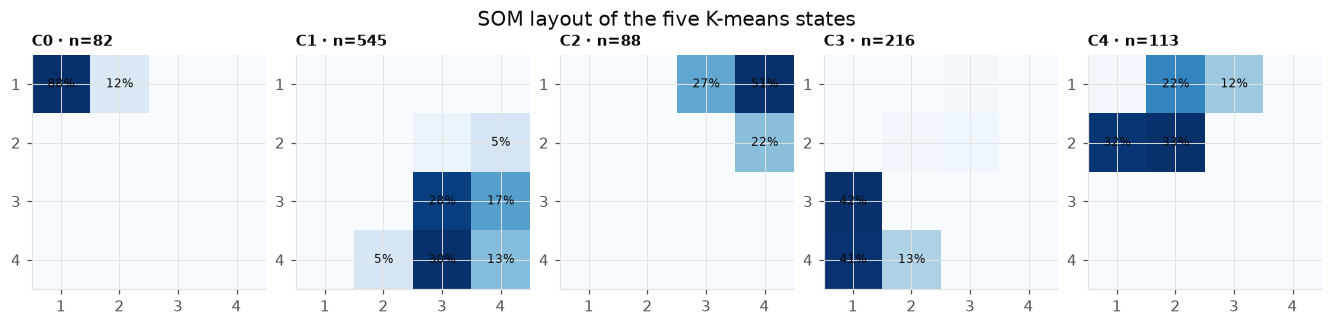

In [85]:
node_order=[f"R{i}C{j}" for i in range(1,5) for j in range(1,5)]
mat=pd.crosstab(w.som_node,w.cluster).reindex(index=node_order,columns=range(5),fill_value=0)
fig,axes=plt.subplots(1,5,figsize=(12,2.8),constrained_layout=True)
for c,ax in enumerate(axes):
    shares=mat[c].to_numpy().reshape(4,4)/mat[c].sum()
    ax.imshow(shares,cmap="Blues",vmin=0,vmax=max(.25,shares.max()))
    ax.set_title(f"C{c} · n={mat[c].sum()}",fontsize=10)
    ax.set_xticks(range(4),[1,2,3,4]);ax.set_yticks(range(4),[1,2,3,4])
    for (i,j),v in np.ndenumerate(shares):
        if v>0.025:ax.text(j,i,f"{v:.0%}",ha="center",va="center",fontsize=8)
fig.suptitle("SOM layout of the five K-means states",fontsize=13)
fig.savefig(OUT/"section9_som_cluster_overlay.png",dpi=200)
plt.show()

**Interpretation.** C0 is concentrated on one node; the much larger C1 occupies a wider part of the grid. Grid position expresses sensor similarity, not clock time or the physical room layout.

### Global IF vs consensus flags

**Question:** Does a global detector treat high-activity readings differently from a state-aware consensus?

In [86]:
ranks=w[["score_iso_global","score_lof","score_centroid","score_iso_state"]].rank(pct=True)
w["global_if"] = ranks.score_iso_global.ge(.95)
w["lof53"] = ranks.score_lof.ge(.95)
votes = ranks[["score_lof","score_centroid","score_iso_state"]].ge(.95).sum(axis=1)
assert votes.eq(w.anomaly_votes).all()
assert votes.ge(2).equals(w.consensus)
assert (w.consensus.sum(),w.global_if.sum(),w.lof53.sum())==(39,53,53)
rates = w.groupby(["cluster","state"])[["consensus","global_if","lof53"]].agg(["sum","mean"])
display(rates.round(3))
print("High-activity IF:",int(w.loc[w.cluster.eq(0),"global_if"].sum()),"of 82 windows")

consensus        global_if        lof53       
                                         sum   mean       sum   mean   sum   mean
cluster state                                                                    
0       High activity                      7  0.085        42  0.512     6  0.073
1       Dark / quiet                      19  0.035         0  0.000    37  0.068
2       Elevated, falling CO₂              3  0.034         0  0.000     1  0.011
3       Illuminated / mostly empty         9  0.042         0  0.000     8  0.037
4       Moderate activity                  1  0.009        11  0.097     1  0.009

High-activity IF: 42 of 82 windows


### Anomaly rate by room state

**Question:** How does knowing the state change which observations deserve review?

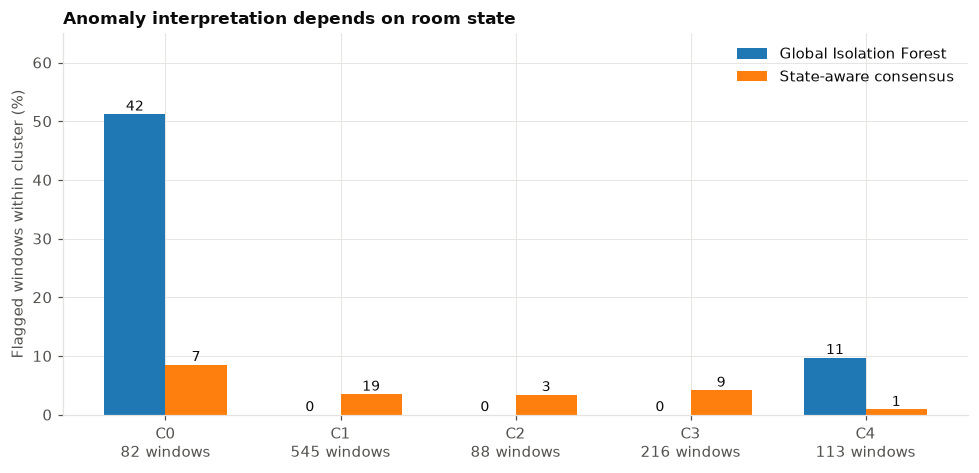

In [87]:
counts=w.groupby("cluster").size().reindex(range(5))
sums=w.groupby("cluster")[["global_if","consensus"]].sum().reindex(range(5))
fig,ax=plt.subplots(figsize=(9,4.4))
x=np.arange(5);width=.35
for shift,field,label in [(-width/2,"global_if","Global Isolation Forest"),(width/2,"consensus","State-aware consensus")]:
    vals=100*sums[field].to_numpy()/counts.to_numpy()
    bars=ax.bar(x+shift,vals,width,label=label)
    for bar,count in zip(bars,sums[field]):
        ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.6,str(count),ha="center",fontsize=9)
ax.set_xticks(x,[f"C{i}\n{counts[i]} windows" for i in range(5)])
ax.set_ylabel("Flagged windows within cluster (%)")
ax.set_title("Anomaly interpretation depends on room state")
ax.legend(frameon=False)
ax.set_ylim(0,65)
fig.tight_layout();fig.savefig(OUT/"section9_anomaly_by_state.png",dpi=220);plt.show()

### Refit K-Means after anomaly removal

**Question:** Do the five states survive if flagged windows are withheld during model fitting?

In [88]:
KARGS=dict(n_clusters=5,n_init=20,random_state=42)
original_labels=w.cluster.to_numpy(int)
with threadpool_limits(limits=1):
    km=KMeans(**KARGS).fit(X)
orig_raw=km.predict(X)
overlap=pd.crosstab(original_labels,orig_raw).reindex(index=range(5),columns=range(5),fill_value=0)
rr,cc=linear_sum_assignment(-overlap.to_numpy())
aligned_map=dict(zip(overlap.columns[cc],overlap.index[rr]))
assert np.array_equal(np.array([aligned_map[i] for i in orig_raw]),original_labels)
reference_centres=np.vstack([km.cluster_centers_[key] for key in [next(k for k,v in aligned_map.items() if v==i) for i in range(5)]])

def refit(mask):
    mask=np.asarray(mask,dtype=bool)
    with threadpool_limits(limits=1): model=KMeans(**KARGS).fit(X[~mask])
    proposed=model.predict(X)
    ct=pd.crosstab(original_labels,proposed).reindex(index=range(5),columns=range(5),fill_value=0)
    i,j=linear_sum_assignment(-ct.to_numpy());mapping=dict(zip(ct.columns[j],ct.index[i]))
    aligned=np.array([mapping[k] for k in proposed])
    centres=np.vstack([model.cluster_centers_[next(k for k,v in mapping.items() if v==i)] for i in range(5)])
    moves=np.linalg.norm(centres-reference_centres,axis=1)
    return {"removed":int(mask.sum()),"changed":int((aligned!=original_labels).sum()),
            "ARI":adjusted_rand_score(original_labels,aligned),
            "largest_centroid_shift":moves.max(),"C0_centroid_shift":moves[0]},aligned

policies={"Consensus":w.consensus.to_numpy(bool),"Global IF":w.global_if.to_numpy(bool),
          "LOF":w.lof53.to_numpy(bool)}
observed={name:refit(mask)[0] for name,mask in policies.items()}
results=pd.DataFrame(observed).T
display(results.round(3))
assert int(results.loc["Consensus","changed"])==11

,removed,changed,ARI,largest_centroid_shift,C0_centroid_shift
Consensus,39.0,11.0,0.977,0.697,0.697
Global IF,53.0,25.0,0.980,2.218,2.218
LOF,53.0,3.0,0.994,0.623,0.623


**Interpretation.** Removing consensus flags changes only 11/1,044 assignments (ARI 0.977). This indicates strong persistence of the five broad states, but does not prove that excluding the readings improves the model.

### Control for ordinary deletion and state imbalance

**Question:** Are anomaly-selected removals more disruptive than random removals?

In [89]:
# Full 500-draw controls are supplied from the executed Investigation 4 notebook.
# Set True to rebuild every refit from the matched 24-feature windows (slow).
RECOMPUTE_ALL_CONTROLS = False
CONTROL_DRAWS = 500
if RECOMPUTE_ALL_CONTROLS:
    seeds=iter(np.random.SeedSequence(4368003).spawn(6))
    state_rows=[np.flatnonzero(original_labels==i) for i in range(5)]
    rows=[]
    for name,mask in policies.items():
        ns=[int(mask[idx].sum()) for idx in state_rows]
        for method in ["Equal-size random","Cluster-stratified random"]:
            rng=np.random.default_rng(next(seeds))
            for draw in range(CONTROL_DRAWS):
                if method=="Equal-size random":
                    chosen=rng.choice(len(w),int(mask.sum()),replace=False)
                else: 
                    chosen=np.concatenate([rng.choice(idx,n,replace=False)
                                           for idx,n in zip(state_rows,ns)])
                selected=np.zeros(len(w),bool);selected[chosen]=True
                metric,_=refit(selected)
                rows.append({"policy":name,"control":method,"draw":draw+1,
                             "changed_all":metric["changed"],
                             "max_centre_shift":metric["largest_centroid_shift"]})
    controls=pd.DataFrame(rows)
else:
    controls=pd.read_csv(ROOT/"evidence/random_removal_all_draws.csv")
    control_check=pd.read_csv(ROOT/"evidence/targeted_removal_effects.csv")
    for label in policies:
        row=control_check.loc[control_check.policy.eq(label)].iloc[0]
        assert int(row.changed_all)==int(results.loc[label,"changed"])
        assert abs(row.ARI_all-results.loc[label,"ARI"])<1e-10
    assert controls.groupby(["policy","control"]).size().eq(CONTROL_DRAWS).all()

summary=controls.groupby(["policy","control"])[["changed_all","max_centre_shift"]].quantile([.025,.5,.975]).round(3)
display(summary)

changed_all  max_centre_shift
policy    control                                                       
Consensus Cluster-stratified random 0.025          0.0             0.118
                                    0.500          1.0             0.191
                                    0.975          9.0             0.315
          Equal-size random         0.025          0.0             0.069
                                    0.500          2.0             0.140
                                    0.975          9.0             0.293
Global IF Cluster-stratified random 0.025          0.0             0.415
                                    0.500          5.0             0.841
                                    0.975         24.0             1.608
          Equal-size random         0.025          0.0             0.089
                                    0.500          2.0             0.173
                                    0.975         10.0             0.322
LOF       Cluster-stratified random 0.025          0.0             0.101
                                    0.500          1.0             0.166
                                    0.975          8.0             0.279
          Equal-size random         0.025          0.0             0.083
                                    0.500          2.0             0.169
                                    0.975         10.0             0.327

### Poster figure: targeted removal versus controls

**Question:** Do the observed membership changes exceed the random-removal reference ranges?

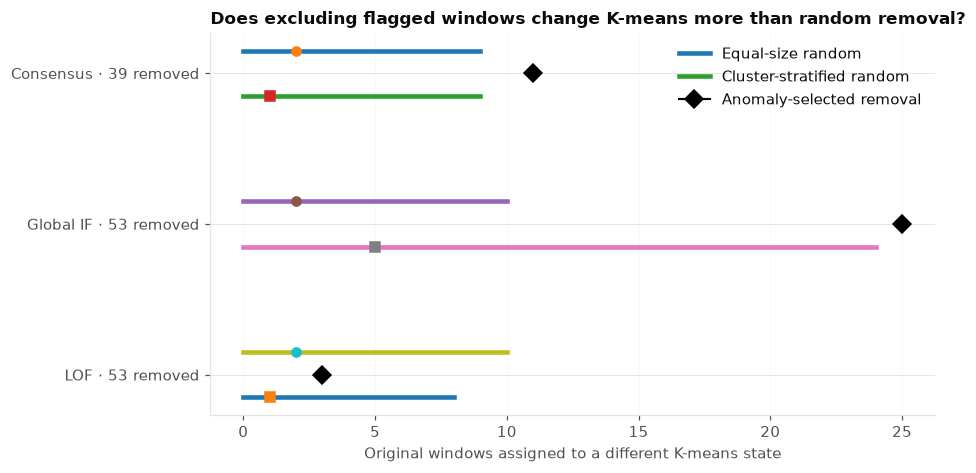

In [90]:
fig,ax=plt.subplots(figsize=(8.7,4.4))
names=list(policies)
for row,name in enumerate(names):
    for delta,kind,marker in [(-.15,"Equal-size random","o"),(.15,"Cluster-stratified random","s")]:
        x=controls.loc[(controls.policy==name)&(controls.control==kind),"changed_all"]
        lo,mid,hi=x.quantile([.025,.5,.975])
        ax.plot([lo,hi],[row+delta]*2,lw=3,label=kind if row==0 else None)
        ax.plot(mid,row+delta,marker=marker,ms=6)
    ax.plot(results.loc[name,"changed"],row,marker="D",color="black",ms=8,
            label="Anomaly-selected removal" if row==0 else None)
ax.set_yticks(range(len(names)),[f"{name} · {int(results.loc[name,'removed'])} removed" for name in names])
ax.invert_yaxis();ax.set_xlabel("Original windows assigned to a different K-means state")
ax.set_title("Does excluding flagged windows change K-means more than random removal?")
ax.legend(frameon=False,loc="upper right");ax.grid(axis="x",alpha=.2)
fig.tight_layout();fig.savefig(OUT/"section9_cluster_removal_controls.png",dpi=220);plt.show()

**Interpretation.** The archived 500-draw controls provide a distribution for each removal policy. The five broad room profiles persist, although individual cases and C0 centroid location can shift.

### Consider recorded and detected events

**Question:** Do anomaly flags plausibly coincide with departures or arrivals?

In [91]:
# Present the checked event-overlap audit, without treating predicted events as ground truth.
events=load("arash/v6_detected_events_with_official_group_clusters.csv")
recorded=pd.read_csv(SOURCE/"arash/ground_truth_room_transitions_EVALUATION_ONLY.csv")
summary=pd.read_csv(ROOT/"evidence/event_overlap_consensus_window_and_episode_denominators.csv")
assert len(recorded)==8
assert len(events)==10
assert int(w.consensus.sum())==int(summary.all_consensus_windows.iloc[0])==39
display(summary[["source","events_with_consensus_within_5min",
                 "unique_consensus_episodes_within_5min","all_consensus_episodes"]])
print("Detected events with official cluster:",int(events.has_group_cluster.sum()),"of",len(events))

,source,events_with_consensus_within_5min,unique_consensus_episodes_within_5min,all_consensus_episodes
0,Detected,1,1,28
1,Recorded,1,1,28


Detected events with official cluster: 9 of 10


**Interpretation.** A consensus-flagged episode occurs near one recorded departure, but overall event/anomaly overlap is consistent with matched recording-time controls. A detected event cannot be treated as independent ground truth for an anomaly.

### Reproducible Section 9 evidence summary

**Question:** Which findings should be reported in the poster and which belong in supporting work?

In [92]:
poster_stats=pd.DataFrame([
    {"result":"Room-state structure","value":"5 K-means states across 1,044 windows"},
    {"result":"Global IF in high activity","value":f"{int(w.loc[w.cluster.eq(0),'global_if'].sum())}/82"},
    {"result":"Avani consensus windows","value":str(int(w.consensus.sum()))},
    {"result":"Consensus-removal membership changes","value":str(int(results.loc['Consensus','changed']))},
    {"result":"Consensus-removal ARI","value":f"{results.loc['Consensus','ARI']:.3f}"},
    {"result":"K-means/GMM ARI","value":f"{adjusted_rand_score(b.cluster,b.label_gmm):.3f}"},
    {"result":"1-min vs 5-min cluster ARI","value":f"{comparison.iloc[0]:.3f}"},
])
display(poster_stats)
poster_stats.to_csv(OUT/"section9_summary.csv",index=False)

,result,value
0,Room-state structure,"5 K-means states across 1,044 windows"
1,Global IF in high activity,42/82
2,Avani consensus windows,39
3,Consensus-removal membership changes,11
4,Consensus-removal ARI,0.977
5,K-means/GMM ARI,0.762
6,1-min vs 5-min cluster ARI,0.854


### conclusion and limitations

Combining clustering with anomaly detection changes what an unusual reading means. Global Isolation Forest selects many high-activity observations that form a coherent occupied state; Avani's consensus highlights a different set of windows across the five states. Excluding the 39 consensus windows changes only 11 K-means assignments, so the broad room-state structure persists, although selected observations can shift cluster centres more than randomly removed data. SOM shows finer variations within the broad states; window-length tests show that exact anomaly-review lists are more sensitive to temporal aggregation than cluster groupings. A departure-related example provides plausible behavioural context, but the small number of recorded transitions does not establish a general event–anomaly link.

**Cautions:** 7 dates, substantial gaps, temporal dependence, unequal state sizes, shared sensor evidence across algorithms, and no confirmed fault labels. A statistical anomaly is not proof of a sensor fault. Maintain the team's original Sections 1–8 and integrate these cells once to avoid duplicating Avani's or Arash's methods.

**AI integrity:** This draft section was prepared with AI assistance from the investigator's verified results and requires group review, attribution, and complete execution in the final shared notebook before submission.

## References
- Singh, A. P., Jain, V., Chaudhari, S., Kraemer, F. A., Werner, S. and Garg, V. (2018) 'Machine learning-based occupancy estimation using multivariate sensor nodes', *2018 IEEE Globecom Workshops (GC Wkshps)*, pp. 1–6.
- Singh, A. P. and Chaudhari, S. (2018) *Room Occupancy Estimation* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5P605